<a href="https://colab.research.google.com/github/Emberits/ice_shedding_app/blob/main/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%22Mak_Gor_v_4_1_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
#старый номер ячейки - 1
# Блок A1 — создание структуры каталогов проекта
import os

base_dir = "/content/hoarfrost_project"
os.makedirs(os.path.join(base_dir, "config"), exist_ok=True)
os.makedirs(os.path.join(base_dir, "src"), exist_ok=True)
os.makedirs(os.path.join(base_dir, "data"), exist_ok=True)
os.makedirs(os.path.join(base_dir, "output"), exist_ok=True)

print("Project directories created under", base_dir)

Project directories created under /content/hoarfrost_project


In [3]:
import os
import shutil
import zipfile

archive = "/content/drive/MyDrive/hoarfrost_project_backups/hoarfrost_project_2026-09-19_4.zip"
local_archive = "/content/hoarfrost_project_2026-09-19_4.zip"
restore_dir = "/content/"

# Копируем архив с Google Drive на локальную ВМ Colab
shutil.copy2(archive, local_archive)

# Создаем папку для восстановленных данных
#os.makedirs(restore_dir, exist_ok=True)

# Распаковываем архив
with zipfile.ZipFile(local_archive, "r") as z:
    z.extractall(restore_dir)

print("Готово:", restore_dir)
!find /content/restored_data -maxdepth 2 -type f | head

Готово: /content/
find: ‘/content/restored_data’: No such file or directory


In [4]:
import sys
import importlib
from pathlib import Path

PROJECT_ROOT = Path("/content/hoarfrost_project")

if not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"Project directory not found: {PROJECT_ROOT}"
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.makkonen_model as makkonen_model
import src.simulation_runner as simulation_runner
import src.calibration as calibration

importlib.reload(makkonen_model)
importlib.reload(simulation_runner)
importlib.reload(calibration)

print("Project root:", PROJECT_ROOT)
print("Makkonen:", makkonen_model.__file__)
print("Runner:", simulation_runner.__file__)
print("Calibration:", calibration.__file__)

Project root: /content/hoarfrost_project
Makkonen: /content/hoarfrost_project/src/makkonen_model.py
Runner: /content/hoarfrost_project/src/simulation_runner.py
Calibration: /content/hoarfrost_project/src/calibration.py


In [5]:
#старый номер ячейки - 2
!pip install pvlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.4/19.4 MB 86.3 MB/s eta 0:00:00


In [ ]:
СТОП

In [6]:
#старый номер ячейки - 3
import numpy as np
import pandas as pd
import pvlib


def compute_qsw_from_pvlib(
    timestamps_utc: pd.Series,
    ntenths: pd.Series,
    lat: float = 62.03389,
    lon: float = 129.73306,
    altitude_m: float = 100.0,
) -> pd.Series:
    """
    Расчёт qSWperm2 (W/m^2) по UTC-времени, координатам и облачности ntenths.
    timestamps_utc: pandas Series или array-like с временем в UTC.
    ntenths: облачность в десятых (0..8).
    """

    # 1. Время -> DatetimeIndex, обязательно tz-aware UTC
    ts = pd.to_datetime(timestamps_utc, errors="coerce")

    if isinstance(ts, pd.Series):
        valid_index = ts.index
        ts_index = pd.DatetimeIndex(ts)
    else:
        valid_index = None
        ts_index = pd.DatetimeIndex(ts)

    if ts_index.tz is None:
        ts_index = ts_index.tz_localize("UTC")
    else:
        ts_index = ts_index.tz_convert("UTC")

    # 2. Облачность
    nt = pd.to_numeric(ntenths, errors="coerce").fillna(0.0).clip(lower=0.0, upper=8.0)

    # 3. Локация
    location = pvlib.location.Location(
        latitude=lat,
        longitude=lon,
        tz="UTC",
        altitude=altitude_m,
        name="Yakutsk",
    )

    # 4. Clear-sky irradiance
    cs = location.get_clearsky(ts_index, model="ineichen")
    ghi_clear = cs["ghi"].astype(float)

    # 5. Ослабление из-за облаков
    cloud_factor = 0.8
    f_cloud = 1.0 - cloud_factor * (nt.to_numpy() / 8.0)
    f_cloud = np.clip(f_cloud, 0.2, 1.0)

    qsw = ghi_clear.to_numpy() * f_cloud

    # 6. Возвращаем Series в том же порядке
    if valid_index is None:
        return pd.Series(qsw)
    return pd.Series(qsw, index=valid_index, name="qSWperm2")

In [15]:
#новая консттанты
%%writefile /content/hoarfrost_project/config/constants.py
# -*- coding: utf-8 -*-
'''
Единый runtime-реестр параметров case_01.

Источники:
- input_case_01_numeric_registry.updated.md;
- variables_case_01_registry.updated.md.

Гипотеза ориентации для Горячева V2:
    phiH_deg  = -ugol2_deg
    phiK1_deg = +ugol1_deg
'''

from __future__ import annotations

from dataclasses import asdict
from typing import Dict

from src.common_types import CableParams


PROJECT_CONSTANTS_VERSION = "1.1.0"
CASE_ID = "case_01"
SPAN_ID = "vl_35_kv"


# Геометрия, механика и электрические параметры case_01.
L_M = 151.0
D_PR_M = 0.0114
F_M2 = 0.00007939

BETA_1_PER_C = 0.0000192
T0_C = 20

A_N = 6542250
B_N_M2 = 4.73
C_N_M = 3.000

#было
#A_N = 6549675.0
#B_N_M2 = 2.331
#C_N_M = 3.998

Q0T_N_PER_M = 2.7
R_OHM_PER_M = 0.0004218

HEIGHT_DIFFERENCE_M = 0.0


# Физические константы.
G_M_PER_S2 = 9.81
SIGMA_W_PER_M2_K4 = 5.670367e-8

CP_J_PER_KG_K = 1000.0
KA_W_PER_M_K = 0.026
LE_J_PER_KG = 2_833_000.0

RHO_C_KG_PER_M3 = 2700.0
C_C_J_PER_KG_K = 920.0


# Общие policy и fallback.
DEFAULT_PRESSURE_PA = 101325.0
FILL_MISSING_WIND_WITH_ZERO = True

RESET_IF_TA_ABOVE_ZERO = True
RESET_IF_T1_ABOVE_ZERO = True

# Горячев: коэффициент формулы (12) должен быть согласован
# с goryachev_model.py и формульным реестром.
GORYACHEV_GRAVITY_M_PER_S2 = 9.81


# Версии данных и pipeline.
DF_NORM_SCHEMA_VERSION = "1.1.0"
DF_CAL_SCHEMA_VERSION = "1.1.0"
DF_SIM_SCHEMA_VERSION = "1.1.0"


# Горячев: mapping углов и сегментная калибровка.
GORYACHEV_ANGLE_MAPPING_VERSION = "hypothesis_v2"
GORYACHEV_REFERENCE_MODE = "segment_no_ice_median"

GORYACHEV_RAW_PHI_H_COLUMN = "ugol2"
GORYACHEV_RAW_PHI_K1_COLUMN = "ugol1"

GORYACHEV_PHI_H_SIGN = -1.0
GORYACHEV_PHI_K1_SIGN = 1.0

GORYACHEV_MIN_REFERENCE_ROWS_PER_MONTH = 20
GORYACHEV_BASELINE_JUMP_THRESHOLD_DEG = 3.0
GORYACHEV_RAW_ANGLE_ABS_LIMIT_DEG = 45.0

GORYACHEV_MIN_SAG_M = 0.01
GORYACHEV_MAX_SAG_M = 100.0
GORYACHEV_MIN_L0_OVER_SPAN = 0.5
GORYACHEV_MAX_L0_OVER_SPAN = 2.0

# ---------------------------------------------------------------------------
# Reviewed raw-angle segmentation for the historical case_01 dataset.
#
# This registry is intentionally case-specific. It must not be interpreted as
# a universal rule for new spans, other sensors, or future time intervals.
#
# (timestamp_start, canonical_segment_id, canonical_segment_role)
# ---------------------------------------------------------------------------

GORYACHEV_ORIENTATION_SEGMENTATION_MODE = (
    "reviewed_case_01"
)

CASE_01_CANONICAL_ANGLE_BOUNDARIES = (
    (
        "2023-12-13 05:43:48",
        1,
        "stable_historical_regime_A",
    ),
    (
        "2025-01-06 04:28:34",
        2,
        "transition_regime_2025",
    ),
    (
        "2025-02-26 05:38:46",
        3,
        "stable_regime_B",
    ),
    (
        "2026-01-01 03:17:07",
        4,
        "stable_post_change_regime_C",
    ),
)


def build_cable_case_01() -> CableParams:
    return CableParams(
        dprm=D_PR_M,
        lm=L_M,
        Fm2=F_M2,
        AN=A_N,
        BNm2=B_N_M2,
        CNm=C_N_M,
        beta1perC=BETA_1_PER_C,
        T0C=T0_C,
        q0TNperm=Q0T_N_PER_M,
        Rohmperm=R_OHM_PER_M,
    )


def alpha_star_case_01() -> float:
    effective_stiffness_n = (
        A_N - C_N_M ** 2 / B_N_M2
    )

    if effective_stiffness_n <= 0.0:
        raise ValueError(
            "Недопустимая эффективная жёсткость: "
            "A_N - C_N_M^2 / B_N_M2 <= 0."
        )

    return 1.0 / effective_stiffness_n


def case_01_constants_report() -> Dict[str, object]:
    cable = build_cable_case_01()

    return {
        "project_constants_version": (
            PROJECT_CONSTANTS_VERSION
        ),
        "case_id": CASE_ID,
        "span_id": SPAN_ID,
        "effective_stiffness_n": (
            A_N - C_N_M ** 2 / B_N_M2
        ),
        "alpha_star_1_per_n": alpha_star_case_01(),
        **asdict(cable),
    }


Overwriting /content/hoarfrost_project/config/constants.py


In [ ]:
#новая консттанты
%%writefile /content/hoarfrost_project/config/__init__.py
# Пакет конфигурации проекта.


In [ ]:
#старый номер ячейки - 4
%%writefile /content/hoarfrost_project/src/common_types.py
# -*- coding: utf-8 -*-

from dataclasses import dataclass
from typing import Optional


@dataclass
class MeteoInput:
    """
    Единый вход метео/тепловых данных для одного шага модели Макконена.

    prevdeltaTcK_init:
        Стартовое значение ΔTc для первого шага расчёта.
        Используется только если в состоянии ещё нет TcprevC/T1prevC.
    """
    taC: float
    T1C: float
    eaPa: float
    paPa: float
    vmpers: float
    ntenths: float
    qSWperm2: float
    QJWperm: float
    deltataus: float
    prevdeltaTcK_init: float = 0.0


@dataclass
class CableParams:
    """
    Параметры провода.

    Для Макконена сейчас обязателен только dprm.
    Остальные поля — задел под Горячева/механику.
    """
    dprm: float
    lm: Optional[float] = None
    Fm2: Optional[float] = None
    AN: Optional[float] = None
    BNm2: Optional[float] = None
    CNm: Optional[float] = None
    beta1perC: Optional[float] = None
    T0C: Optional[float] = None
    q0TNperm: Optional[float] = None
    Rohmperm: Optional[float] = None


@dataclass
class HoarfrostState:
    """
    Состояние изморози/инея на текущем шаге.

    TcprevC:
        Предыдущее расчётное значение температуры кабеля (Tc) из Макконена.
    T1prevC:
        Предыдущее измеренное значение температуры оболочки T1 из данных.
    prevdeltaTcK:
        ΔTc, использованная на прошлом шаге в уравнении переходного теплового потока.
    """
    Hm: float = 0.0
    rhotkgm3: float = 0.0
    masspermkgm: float = 0.0
    prevdeltaTcK: float = 0.0
    TcprevC: Optional[float] = None
    T1prevC: Optional[float] = None


@dataclass
class GoryachevCalibrationParams:
    """
    Калибровочные параметры для механического слоя (Горячев).
    """
    TcalC: float
    phiHcaldeg: float
    phiK1caldeg: float


@dataclass
class MechanicalState:
    """
    Состояние/диагностика механического слоя.
    """
    q0gkgm3: Optional[float] = None
    L0g: Optional[float] = None
    FgN: Optional[float] = None
    cgoryachevm: Optional[float] = None


@dataclass
class CoupledState:
    """
    Совмещённое состояние для интеграции Макконен + Горячев.
    """
    hoarfrost: HoarfrostState
    mechanical: Optional[MechanicalState] = None


In [ ]:
%%writefile /content/hoarfrost_project/src/data_normalization.py
# -*- coding: utf-8 -*-
"""
data_normalization.py
=====================

Единый модуль подготовки входов для модели изморози.

Содержит:
- чтение исходных CSV;
- выбор единственного источника тока:
  No0036 positive event-state hold -> No0039 fallback;
- backward merge No0039 и Meteostation;
- лимит давности Meteostation;
- явные policies пропусков;
- формирование канонической схемы;
- audit/provenance.

Канонические единицы:
- Ta_C, T1_C: °C;
- wind_m_s: m/s;
- pressure_Pa, vapor_pressure_Pa: Pa;
- cloud_tenths: tenths;
- solar_W_m2: W/m²;
- current_A: A.

Ток выбирается один раз и далее не изменяется.

Meteo age policy:
- прошлое измерение Meteostation можно применять не более 3 часов;
- если wind отсутствует/устарел: wind_m_s = 0.0;
- если pressure отсутствует/устарел: pressure_Pa = 101325.0;
- все такие строки помечаются quality/provenance fields.
"""

from __future__ import annotations

from dataclasses import dataclass, field
from pathlib import Path
from typing import Any, Dict, Iterable, Optional, Sequence

import numpy as np
import pandas as pd


# ---------------------------------------------------------------------------
# Global policies
# ---------------------------------------------------------------------------

CURRENT_POLICY_NAME = (
    "No0036_positive_event_hold_then_"
    "No0039_fallback_no_postprocessing"
)

DEFAULT_CURRENT_A = 0.0

METEO_MAX_AGE_SECONDS = 3 * 60 * 60
DEFAULT_WIND_M_S = 0.0
DEFAULT_PRESSURE_PA = 101325.0

CANONICAL_COLUMNS: tuple[str, ...] = (
    "timestamp",
    "Ta_C",
    "T1_C",
    "wind_m_s",
    "pressure_Pa",
    "vapor_pressure_Pa",
    "cloud_tenths",
    "solar_W_m2",
    "current_A",
)

REQUIRED_CANONICAL_COLUMNS: tuple[str, ...] = (
    "timestamp",
    "Ta_C",
    "T1_C",
    "wind_m_s",
    "pressure_Pa",
    "vapor_pressure_Pa",
    "current_A",
)

CURRENT_SOURCE_PRIORITY: tuple[str, ...] = (
    "current_A",
    "current_a",
    "I_A",
    "i_A",
    "I",
    "i",
    "current",
    "ток_А",
    "ток_а",
    "ток",
    "Ток, А",
    "Ток А",
)

COLUMN_ALIASES: Dict[str, tuple[str, ...]] = {
    "timestamp": (
        "timestamp",
        "datetime",
        "date_time",
        "date",
        "time",
        "created_at",
        "Дата",
        "дата",
        "Дата/время",
        "Дата и время",
        "Время",
    ),
    "Ta_C": (
        "Ta_C",
        "taC",
        "ta_c",
        "Ta",
        "ta",
        "air_temperature_C",
        "air_temp_C",
        "temperature_C",
        "tvozd",
        "Температура воздуха, °C",
        "Температура воздуха",
        "Температура, °C",
    ),
    "T1_C": (
        "T1_C",
        "t1C",
        "t1_c",
        "T1",
        "t1",
        "tcab",
        "conductor_temperature_C",
        "wire_temperature_C",
        "cable_temperature_C",
        "Температура провода, °C",
        "Температура провода",
    ),
    "wind_m_s": (
        "wind_m_s",
        "wind_speed_m_s",
        "windspeed2min",
        "aver_speed_10m (fromDB)",
        "wind",
        "Wind",
        "v",
        "V",
        "Скорость ветра, м/с",
        "Скорость ветра",
    ),
    "pressure_Pa": (
        "pressure_Pa",
        "pressure_pa",
        "p_Pa",
        "pressureGPa",
        "p",
        "P",
        "pressure",
        "Давление, Па",
        "Давление, hPa",
        "Давление, гПа",
    ),
    "vapor_pressure_Pa": (
        "vapor_pressure_Pa",
        "vapour_pressure_Pa",
        "ea_Pa",
        "ea",
        "e_a",
        "e",
        "vapor_pressure",
        "Парциальное давление пара, Па",
    ),
    "cloud_tenths": (
        "cloud_tenths",
        "cloudiness_tenths",
        "cloud",
        "cloudiness",
        "n",
        "N",
        "Облачность",
    ),
    "solar_W_m2": (
        "solar_W_m2",
        "solar",
        "solar_radiation",
        "shortwave_W_m2",
        "qSW",
        "qsw",
        "Солнечная радиация, Вт/м2",
        "Солнечная радиация, Вт/м²",
    ),
    "current_A": CURRENT_SOURCE_PRIORITY,
}


# ---------------------------------------------------------------------------
# Configuration and result containers
# ---------------------------------------------------------------------------

@dataclass(frozen=True)
class SourceFileConfig:
    sensor_main_time_column: str = "created_at"
    sensor_current_time_column: str = "created_at"
    primary_current_column: str = "iideistv"
    auxiliary_current_column: str = "iideistv"
    meteo_time_column: str = "created_at"
    max_meteo_age_seconds: int = METEO_MAX_AGE_SECONDS
    default_wind_m_s: float = DEFAULT_WIND_M_S
    default_pressure_pa: float = DEFAULT_PRESSURE_PA


@dataclass
class NormalizationResult:
    dataframe: pd.DataFrame
    provenance: Dict[str, Any] = field(
        default_factory=dict
    )

    def copy(self) -> "NormalizationResult":
        return NormalizationResult(
            dataframe=self.dataframe.copy(),
            provenance=dict(self.provenance),
        )


# ---------------------------------------------------------------------------
# Generic helpers
# ---------------------------------------------------------------------------

def _normalise_column_name(
    name: object,
) -> str:
    return (
        str(name)
        .strip()
        .replace("\n", " ")
        .replace("\xa0", " ")
        .casefold()
    )


def _column_lookup(
    columns: Iterable[object],
) -> Dict[str, str]:
    lookup: Dict[str, str] = {}

    for column in columns:
        normalised = _normalise_column_name(
            column
        )

        if normalised not in lookup:
            lookup[normalised] = str(column)

    return lookup


def find_column(
    dataframe: pd.DataFrame,
    candidates: Sequence[str],
) -> Optional[str]:
    lookup = _column_lookup(
        dataframe.columns
    )

    for candidate in candidates:
        normalised_candidate = _normalise_column_name(
            candidate
        )

        if normalised_candidate in lookup:
            return lookup[normalised_candidate]

    return None


def _first_present_column(
    dataframe: pd.DataFrame,
    candidates: Sequence[str],
) -> Optional[str]:
    for candidate in candidates:
        if candidate in dataframe.columns:
            return candidate

    return None


def _coerce_numeric(
    series: pd.Series,
) -> pd.Series:
    if pd.api.types.is_numeric_dtype(series):
        return pd.to_numeric(
            series,
            errors="coerce",
        )

    prepared = (
        series.astype("string")
        .str.strip()
        .str.replace("\u2212", "-", regex=False)
        .str.replace(",", ".", regex=False)
        .str.replace(r"\s+", "", regex=True)
    )

    return pd.to_numeric(
        prepared,
        errors="coerce",
    )


def _normalise_timestamp(
    series: pd.Series,
) -> pd.Series:
    """
    Parses timestamps without warning on ISO8601 strings.

    Order:
    1. already datetime64;
    2. ISO8601 strings, e.g. YYYY-MM-DD HH:MM:SS;
    3. day-first fallback for formats such as DD.MM.YYYY HH:MM.
    """
    if pd.api.types.is_datetime64_any_dtype(
        series
    ):
        return pd.to_datetime(
            series,
            errors="coerce",
        )

    as_text = series.astype("string")

    parsed = pd.to_datetime(
        as_text,
        errors="coerce",
        format="ISO8601",
    )

    unresolved = parsed.isna() & as_text.notna()

    if bool(unresolved.any()):
        parsed_fallback = pd.to_datetime(
            as_text.loc[unresolved],
            errors="coerce",
            dayfirst=True,
        )

        parsed.loc[unresolved] = parsed_fallback

    return parsed


def _series_from_column_or_nan(
    dataframe: pd.DataFrame,
    column_name: Optional[str],
) -> pd.Series:
    if column_name is None:
        return pd.Series(
            np.nan,
            index=dataframe.index,
            dtype=float,
        )

    return _coerce_numeric(
        dataframe[column_name]
    )


def _require_columns(
    dataframe: pd.DataFrame,
    columns: Sequence[str],
    dataframe_name: str,
) -> None:
    missing = [
        column
        for column in columns
        if column not in dataframe.columns
    ]

    if missing:
        raise KeyError(
            f"{dataframe_name} is missing "
            f"required columns: {missing}. "
            f"Available columns: "
            f"{list(dataframe.columns)}"
        )


def saturation_vapor_pressure_water_pa(
    temperature_C: pd.Series | float,
) -> pd.Series | float:
    return 611.2 * np.exp(
        17.67
        * temperature_C
        / (
            243.5
            + temperature_C
        )
    )


# ---------------------------------------------------------------------------
# CSV reader
# ---------------------------------------------------------------------------

def read_csv_auto(
    path: str | Path,
) -> pd.DataFrame:
    """
    Читает CSV с распространенными encoding/separator combinations.

    Возвращает dataframe только если разобрано более одной колонки.
    """
    file_path = Path(path)

    if not file_path.exists():
        raise FileNotFoundError(
            f"Input file not found: {file_path}"
        )

    attempts: list[str] = []

    combinations = [
        ("utf-8", ","),
        ("utf-8-sig", ","),
        ("cp1251", ";"),
        ("cp1251", ","),
        ("utf-8", ";"),
        ("utf-8-sig", ";"),
    ]

    for encoding, separator in combinations:
        try:
            dataframe = pd.read_csv(
                file_path,
                encoding=encoding,
                sep=separator,
                low_memory=False,
            )

            if dataframe.shape[1] > 1:
                dataframe.attrs[
                    "csv_encoding"
                ] = encoding

                dataframe.attrs[
                    "csv_separator"
                ] = separator

                return dataframe

            attempts.append(
                f"{encoding}/{separator!r}: "
                f"{dataframe.shape[1]} column"
            )

        except Exception as exc:
            attempts.append(
                f"{encoding}/{separator!r}: "
                f"{type(exc).__name__}: {exc}"
            )

    raise RuntimeError(
        "Could not read CSV file: "
        f"{file_path}\n"
        + "\n".join(attempts)
    )


# ---------------------------------------------------------------------------
# Current source policy
# ---------------------------------------------------------------------------

def _infer_current_unit(
    values: pd.Series,
    source_column: str,
) -> str:
    source_name = _normalise_column_name(
        source_column
    )

    if "ka" in source_name or "ка" in source_name:
        return "kA"

    if (
        "amp" in source_name
        or "а" in source_name
        or source_name in {
            "i",
            "current",
            "ток",
            "current_a",
        }
    ):
        return "A"

    finite_values = values[
        np.isfinite(values)
    ]

    if finite_values.empty:
        return "A"

    max_abs = float(
        finite_values.abs().max()
    )

    if max_abs <= 20.0:
        return "kA"

    return "A"


def _convert_current_to_a(
    values: pd.Series,
    source_column: str,
) -> tuple[pd.Series, str, str]:
    source_unit = _infer_current_unit(
        values,
        source_column,
    )

    if source_unit == "A":
        return (
            values.astype(float),
            source_unit,
            "A_to_A",
        )

    if source_unit == "kA":
        return (
            values.astype(float) * 1000.0,
            source_unit,
            "kA_to_A",
        )

    raise ValueError(
        "Unsupported current unit: "
        f"{source_unit}"
    )


def resolve_current_source(
    dataframe: pd.DataFrame,
    current_source_column: Optional[str] = None,
    default_current_A: float = DEFAULT_CURRENT_A,
) -> tuple[pd.Series, Dict[str, Any]]:
    """
    Generic current resolver.

    Для основного pipeline используйте source-file builder ниже:
    там политика No0036 -> No0039 полностью фиксирована.

    Эта функция сохранена для backward compatibility.
    """
    if current_source_column is not None:
        if current_source_column not in dataframe.columns:
            raise KeyError(
                "Explicit current source column "
                "was not found: "
                f"{current_source_column}"
            )

        source_column = current_source_column
        source_selection = "explicit"

    else:
        source_column = find_column(
            dataframe,
            CURRENT_SOURCE_PRIORITY,
        )

        source_selection = "priority_search"

    if source_column is None:
        values = pd.Series(
            float(default_current_A),
            index=dataframe.index,
            dtype=float,
        )

        return values, {
            "current_policy": (
                "generic_default_constant"
            ),
            "current_source_column": None,
            "current_source_selection": (
                "default_constant"
            ),
            "current_source_unit": "A",
            "current_conversion": "none",
            "current_default_A": float(
                default_current_A
            ),
            "current_missing_count_before_fill": 0,
            "current_missing_count_after_fill": 0,
            "current_postprocessing_applied": False,
            "current_values_modified_after_resolution": (
                False
            ),
        }

    raw_values = _coerce_numeric(
        dataframe[source_column]
    )

    converted_values, source_unit, conversion = (
        _convert_current_to_a(
            raw_values,
            source_column,
        )
    )

    missing_before_fill = int(
        converted_values.isna().sum()
    )

    values = converted_values.fillna(
        float(default_current_A)
    )

    return values.astype(float), {
        "current_policy": (
            "single_explicit_source_no_"
            "postprocessing"
        ),
        "current_source_column": source_column,
        "current_source_selection": (
            source_selection
        ),
        "current_source_unit": source_unit,
        "current_conversion": conversion,
        "current_default_A": float(
            default_current_A
        ),
        "current_missing_count_before_fill": (
            missing_before_fill
        ),
        "current_missing_count_after_fill": int(
            values.isna().sum()
        ),
        "current_postprocessing_applied": False,
        "current_values_modified_after_resolution": (
            False
        ),
    }


def get_current_provenance(
    dataframe: pd.DataFrame,
    current_source_column: Optional[str] = None,
    default_current_A: float = DEFAULT_CURRENT_A,
) -> Dict[str, Any]:
    _, provenance = resolve_current_source(
        dataframe=dataframe,
        current_source_column=current_source_column,
        default_current_A=default_current_A,
    )

    return provenance


def resolve_no0036_no0039_current(
    sensor_main_raw: pd.DataFrame,
    sensor_current_raw: pd.DataFrame,
    config: SourceFileConfig,
) -> tuple[pd.DataFrame, Dict[str, Any]]:
    """
    Creates one explicit current_A field for the No0039 timeline.

    Rule:
    1. Last No0036 event state if value > 0 A.
    2. Otherwise current No0039 value.
    3. Fail if both are unavailable.

    merge_asof(direction="backward") prohibits future current values.
    """
    _require_columns(
        sensor_main_raw,
        [config.sensor_main_time_column],
        "sensor_main_raw",
    )

    _require_columns(
        sensor_current_raw,
        [
            config.sensor_current_time_column,
            config.auxiliary_current_column,
        ],
        "sensor_current_raw",
    )

    sensor_main = sensor_main_raw.copy()
    sensor_auxiliary = sensor_current_raw.copy()

    sensor_main["_sensor_timestamp"] = (
        _normalise_timestamp(
            sensor_main[
                config.sensor_main_time_column
            ]
        )
    )

    sensor_auxiliary["_auxiliary_timestamp"] = (
        _normalise_timestamp(
            sensor_auxiliary[
                config.sensor_current_time_column
            ]
        )
    )

    sensor_main["current_A_primary_0039"] = (
        _coerce_numeric(
            sensor_main.get(
                config.primary_current_column,
                pd.Series(
                    np.nan,
                    index=sensor_main.index,
                ),
            )
        )
    )

    sensor_auxiliary[
        "current_A_auxiliary_0036"
    ] = _coerce_numeric(
        sensor_auxiliary[
            config.auxiliary_current_column
        ]
    )

    sensor_main = (
        sensor_main
        .dropna(
            subset=[
                "_sensor_timestamp",
            ]
        )
        .sort_values("_sensor_timestamp")
        .copy()
    )

    auxiliary_events = (
        sensor_auxiliary
        .dropna(
            subset=[
                "_auxiliary_timestamp",
                "current_A_auxiliary_0036",
            ]
        )
        [
            [
                "_auxiliary_timestamp",
                "current_A_auxiliary_0036",
            ]
        ]
        .rename(
            columns={
                "_auxiliary_timestamp": (
                    "current_A_auxiliary_event_timestamp"
                ),
            }
        )
        .sort_values(
            "current_A_auxiliary_event_timestamp"
        )
        .drop_duplicates(
            subset=[
                "current_A_auxiliary_event_timestamp",
            ],
            keep="last",
        )
        .reset_index(drop=True)
    )

    if auxiliary_events.empty:
        raise RuntimeError(
            "No valid No0036 current events "
            "were found."
        )

    resolved = pd.merge_asof(
        sensor_main,
        auxiliary_events,
        left_on="_sensor_timestamp",
        right_on=(
            "current_A_auxiliary_event_timestamp"
        ),
        direction="backward",
    )

    resolved[
        "current_A_auxiliary_age_seconds"
    ] = (
        resolved["_sensor_timestamp"]
        - resolved[
            "current_A_auxiliary_event_timestamp"
        ]
    ).dt.total_seconds()

    resolved[
        "current_A_from_auxiliary_0036"
    ] = (
        resolved[
            "current_A_auxiliary_0036"
        ].notna()
        & (
            resolved[
                "current_A_auxiliary_0036"
            ]
            > 0.0
        )
    )

    resolved[
        "current_A_from_primary_0039"
    ] = (
        ~resolved[
            "current_A_from_auxiliary_0036"
        ]
        & resolved[
            "current_A_primary_0039"
        ].notna()
    )

    resolved[
        "current_A_missing_after_fallback"
    ] = (
        ~resolved[
            "current_A_from_auxiliary_0036"
        ]
        & ~resolved[
            "current_A_from_primary_0039"
        ]
    )

    resolved[
        "current_A_auxiliary_event"
    ] = (
        resolved[
            "current_A_from_auxiliary_0036"
        ]
        & (
            resolved[
                "current_A_auxiliary_age_seconds"
            ]
            == 0.0
        )
    )

    resolved[
        "current_A_auxiliary_held"
    ] = (
        resolved[
            "current_A_from_auxiliary_0036"
        ]
        & (
            resolved[
                "current_A_auxiliary_age_seconds"
            ]
            > 0.0
        )
    )

    resolved["current_A_source"] = np.select(
        [
            resolved[
                "current_A_auxiliary_event"
            ],
            resolved[
                "current_A_auxiliary_held"
            ],
            resolved[
                "current_A_from_primary_0039"
            ],
        ],
        [
            "auxiliary_0036_event",
            "auxiliary_0036_held",
            "primary_0039_fallback",
        ],
        default="missing_no_current_source",
    )

    resolved["current_A"] = np.where(
        resolved[
            "current_A_from_auxiliary_0036"
        ],
        resolved[
            "current_A_auxiliary_0036"
        ],
        resolved[
            "current_A_primary_0039"
        ],
    )

    partition_columns = [
        "current_A_from_auxiliary_0036",
        "current_A_from_primary_0039",
        "current_A_missing_after_fallback",
    ]

    partition_count = (
        resolved[partition_columns]
        .astype(bool)
        .astype(int)
        .sum(axis=1)
    )

    invalid_partition_rows = int(
        (partition_count != 1).sum()
    )

    if invalid_partition_rows > 0:
        raise RuntimeError(
            "Current-source partition failed: "
            f"{invalid_partition_rows} rows "
            "are not assigned exactly once."
        )

    missing_current_rows = int(
        resolved[
            "current_A_missing_after_fallback"
        ].sum()
    )

    if missing_current_rows > 0:
        raise ValueError(
            "Final current_A missing after "
            "No0036 -> No0039 fallback: "
            f"rows={missing_current_rows}."
        )

    resolved["current_A"] = _coerce_numeric(
        resolved["current_A"]
    )

    if resolved["current_A"].isna().any():
        raise ValueError(
            "current_A contains non-numeric "
            "values after selection."
        )

    if (resolved["current_A"] < 0.0).any():
        raise ValueError(
            "current_A contains negative values "
            "after selection."
        )

    provenance = {
        "current_policy": CURRENT_POLICY_NAME,
        "current_source_column": "current_A",
        "current_source_selection": (
            "explicit_No0036_then_No0039"
        ),
        "current_source_unit": "A",
        "current_conversion": "A_to_A",
        "current_postprocessing_applied": False,
        "current_values_modified_after_resolution": (
            False
        ),
        "current_source_partition_valid": True,
        "n_rows_current_timeline": int(
            len(resolved)
        ),
        "n_auxiliary_0036_rows": int(
            resolved[
                "current_A_from_auxiliary_0036"
            ].sum()
        ),
        "n_auxiliary_0036_event_rows": int(
            resolved[
                "current_A_auxiliary_event"
            ].sum()
        ),
        "n_auxiliary_0036_held_rows": int(
            resolved[
                "current_A_auxiliary_held"
            ].sum()
        ),
        "n_primary_0039_fallback_rows": int(
            resolved[
                "current_A_from_primary_0039"
            ].sum()
        ),
        "n_missing_current_rows": missing_current_rows,
    }

    return resolved, provenance


# ---------------------------------------------------------------------------
# Meteo merge and canonical field construction
# ---------------------------------------------------------------------------

def merge_meteo_on_sensor_timeline(
    sensor_current_resolved: pd.DataFrame,
    meteo_raw: pd.DataFrame,
    config: SourceFileConfig,
) -> tuple[pd.DataFrame, Dict[str, Any]]:
    """
    Backward merges Meteostation onto No0039 timeline.

    The merge itself uses no tolerance so the meteo timestamp and its
    age remain inspectable. Field-level policy later applies the explicit
    max age threshold.
    """
    _require_columns(
        sensor_current_resolved,
        ["_sensor_timestamp"],
        "sensor_current_resolved",
    )

    _require_columns(
        meteo_raw,
        [config.meteo_time_column],
        "meteo_raw",
    )

    meteo = meteo_raw.copy()

    meteo["_meteo_timestamp"] = _normalise_timestamp(
        meteo[
            config.meteo_time_column
        ]
    )

    meteo = (
        meteo
        .dropna(
            subset=[
                "_meteo_timestamp",
            ]
        )
        .sort_values("_meteo_timestamp")
        .drop_duplicates(
            subset=[
                "_meteo_timestamp",
            ],
            keep="last",
        )
        .copy()
    )

    sensor = (
        sensor_current_resolved
        .sort_values("_sensor_timestamp")
        .copy()
    )

    meteo_columns_to_add = [
        column
        for column in meteo.columns
        if column not in sensor.columns
        and column not in {
            config.meteo_time_column,
            "_meteo_timestamp",
        }
    ]

    meteo_right = meteo[
        [
            "_meteo_timestamp",
            *meteo_columns_to_add,
        ]
    ].copy()

    if not meteo_right.columns.is_unique:
        duplicate_columns = (
            meteo_right.columns[
                meteo_right.columns.duplicated()
            ]
            .tolist()
        )

        raise RuntimeError(
            "Meteo merge table has duplicate "
            f"columns: {duplicate_columns}"
        )

    merged = pd.merge_asof(
        sensor,
        meteo_right,
        left_on="_sensor_timestamp",
        right_on="_meteo_timestamp",
        direction="backward",
    )

    merged["timestamp"] = merged[
        "_sensor_timestamp"
    ]

    merged["meteo_age_seconds"] = (
        merged["_sensor_timestamp"]
        - merged["_meteo_timestamp"]
    ).dt.total_seconds()

    merged["meteo_match_found"] = (
        merged["_meteo_timestamp"]
        .notna()
    )

    merged["meteo_age_within_limit"] = (
        merged["meteo_match_found"]
        & (
            merged["meteo_age_seconds"]
            >= 0.0
        )
        & (
            merged["meteo_age_seconds"]
            <= float(
                config.max_meteo_age_seconds
            )
        )
    )

    provenance = {
        "meteo_merge_direction": "backward",
        "meteo_max_age_seconds": int(
            config.max_meteo_age_seconds
        ),
        "meteo_max_age_hours": (
            float(
                config.max_meteo_age_seconds
            )
            / 3600.0
        ),
        "n_sensor_rows": int(len(merged)),
        "n_meteo_matched_rows": int(
            merged["meteo_match_found"].sum()
        ),
        "n_meteo_missing_rows": int(
            (~merged["meteo_match_found"]).sum()
        ),
        "n_meteo_within_age_limit_rows": int(
            merged[
                "meteo_age_within_limit"
            ].sum()
        ),
        "n_meteo_over_age_limit_rows": int(
            (
                merged["meteo_match_found"]
                & ~merged[
                    "meteo_age_within_limit"
                ]
            ).sum()
        ),
    }

    return merged, provenance


def _pressure_to_pa_from_sources(
    dataframe: pd.DataFrame,
) -> tuple[pd.Series, Dict[str, Optional[str]]]:
    direct_pa_column = _first_present_column(
        dataframe,
        [
            "pressure_Pa",
        ],
    )

    hpa_column = _first_present_column(
        dataframe,
        [
            "pressureGPa",
            "pressure_hPa",
            "pressure_hpa",
        ],
    )

    mmhg_column = _first_present_column(
        dataframe,
        [
            "pressuremmHg",
            "press_mm (fromDB)",
            "pressmm",
            "pressure_mmHg",
        ],
    )

    direct_pa = _series_from_column_or_nan(
        dataframe,
        direct_pa_column,
    )

    hpa = _series_from_column_or_nan(
        dataframe,
        hpa_column,
    )

    mmhg = _series_from_column_or_nan(
        dataframe,
        mmhg_column,
    )

    pressure_pa = direct_pa.where(
        direct_pa > 2000.0
    )

    pressure_pa = pressure_pa.fillna(
        hpa.where(
            hpa > 0.0
        ) * 100.0
    )

    pressure_pa = pressure_pa.fillna(
        mmhg.where(
            mmhg > 0.0
        ) * 133.32236842105263
    )

    return pressure_pa, {
        "pressure_direct_pa": direct_pa_column,
        "pressure_hpa": hpa_column,
        "pressure_mmhg": mmhg_column,
    }


def build_canonical_meteo_fields(
    merged_input: pd.DataFrame,
    config: SourceFileConfig,
) -> tuple[pd.DataFrame, Dict[str, Any]]:
    """
    Adds explicit canonical fields to merged raw data.

    Meteo values are accepted only when meteo_age_within_limit is true.
    This is deliberately separate from ffill: the source row timestamp,
    not only field NaN status, controls validity.
    """
    dataframe = merged_input.copy()

    if "timestamp" not in dataframe.columns:
        dataframe["timestamp"] = dataframe[
            "_sensor_timestamp"
        ]

    if "meteo_age_within_limit" not in dataframe.columns:
        raise KeyError(
            "Expected meteo_age_within_limit "
            "after merge_meteo_on_sensor_timeline."
        )

    meteo_valid = dataframe[
        "meteo_age_within_limit"
    ].fillna(False).astype(bool)

    sensor_tcab_column = _first_present_column(
        dataframe,
        [
            "tcab",
            "T1_C",
            "T1C",
        ],
    )

    sensor_tvozd_column = _first_present_column(
        dataframe,
        [
            "tvozd",
            "Ta_C",
            "taC",
        ],
    )

    meteo_temperature_column = _first_present_column(
        dataframe,
        [
            "temperature",
            "temp (fromDB)",
            "temp",
        ],
    )

    sensor_rh_column = _first_present_column(
        dataframe,
        [
            "rh",
            "RH_pct",
            "rhpct",
        ],
    )

    meteo_rh_column = _first_present_column(
        dataframe,
        [
            "humidity",
            "humidity (fromDB)",
        ],
    )

    meteo_wind_column = _first_present_column(
        dataframe,
        [
            "windspeed2min",
            "aver_speed_10m (fromDB)",
            "windmaxspeed2min",
        ],
    )

    T1_sensor_C = _series_from_column_or_nan(
        dataframe,
        sensor_tcab_column,
    )

    Ta_sensor_C = _series_from_column_or_nan(
        dataframe,
        sensor_tvozd_column,
    )

    Ta_meteo_C = _series_from_column_or_nan(
        dataframe,
        meteo_temperature_column,
    )

    RH_sensor_pct = _series_from_column_or_nan(
        dataframe,
        sensor_rh_column,
    )

    RH_meteo_pct = _series_from_column_or_nan(
        dataframe,
        meteo_rh_column,
    )

    raw_wind_m_s = _series_from_column_or_nan(
        dataframe,
        meteo_wind_column,
    ).clip(lower=0.0)

    raw_pressure_Pa, pressure_sources = (
        _pressure_to_pa_from_sources(
            dataframe
        )
    )

    dataframe["T1_C"] = T1_sensor_C

    dataframe["Ta_C"] = Ta_sensor_C.fillna(
        Ta_meteo_C.where(meteo_valid)
    )

    dataframe["RH_pct"] = RH_sensor_pct.fillna(
        RH_meteo_pct.where(meteo_valid)
    ).clip(
        lower=0.0,
        upper=100.0,
    )

    wind_eligible = raw_wind_m_s.where(
        meteo_valid
    )

    pressure_eligible = raw_pressure_Pa.where(
        meteo_valid
    )

    dataframe["wind_m_s_raw"] = raw_wind_m_s
    dataframe["pressure_Pa_raw"] = raw_pressure_Pa

    dataframe["wind_m_s_meteo_valid"] = (
        wind_eligible.notna()
    )

    dataframe["pressure_Pa_meteo_valid"] = (
        pressure_eligible.notna()
    )

    dataframe["wind_m_s"] = wind_eligible.fillna(
        float(config.default_wind_m_s)
    )

    dataframe["pressure_Pa"] = pressure_eligible.fillna(
        float(config.default_pressure_pa)
    )

    dataframe["wind_m_s_defaulted"] = (
        ~dataframe[
            "wind_m_s_meteo_valid"
        ]
    )

    dataframe["pressure_Pa_defaulted"] = (
        ~dataframe[
            "pressure_Pa_meteo_valid"
        ]
    )

    dataframe["vapor_pressure_Pa"] = (
        dataframe["RH_pct"]
        / 100.0
        * saturation_vapor_pressure_water_pa(
            dataframe["Ta_C"]
        )
    )

    dataframe["cloud_tenths"] = 0.0
    dataframe["solar_W_m2"] = 0.0

    dataframe["meteo_quality_status"] = np.select(
        [
            (
                dataframe["wind_m_s_meteo_valid"]
                & dataframe[
                    "pressure_Pa_meteo_valid"
                ]
            ),
            (
                dataframe[
                    "wind_m_s_defaulted"
                ]
                & dataframe[
                    "pressure_Pa_defaulted"
                ]
            ),
            dataframe["wind_m_s_defaulted"],
            dataframe["pressure_Pa_defaulted"],
        ],
        [
            "meteo_valid",
            "wind_and_pressure_defaulted",
            "wind_defaulted",
            "pressure_defaulted",
        ],
        default="meteo_unknown",
    )

    source_report: Dict[
        str,
        Any,
    ] = {
        "T1_C": sensor_tcab_column,
        "Ta_sensor_C": sensor_tvozd_column,
        "Ta_meteo_C": meteo_temperature_column,
        "RH_sensor_pct": sensor_rh_column,
        "RH_meteo_pct": meteo_rh_column,
        "wind_m_s": meteo_wind_column,
        "pressure_sources": pressure_sources,
        "wind_missing_policy": (
            "default_zero_if_missing_or_"
            "meteo_age_exceeds_3h"
        ),
        "pressure_missing_policy": (
            "default_101325Pa_if_missing_or_"
            "meteo_age_exceeds_3h"
        ),
        "cloud_source": (
            "temporary_zero_no_metar_merge"
        ),
        "solar_source": (
            "temporary_zero_no_pvlib"
        ),
        "n_wind_defaulted": int(
            dataframe[
                "wind_m_s_defaulted"
            ].sum()
        ),
        "n_pressure_defaulted": int(
            dataframe[
                "pressure_Pa_defaulted"
            ].sum()
        ),
        "n_meteo_valid": int(
            (
                dataframe[
                    "meteo_quality_status"
                ]
                == "meteo_valid"
            ).sum()
        ),
    }

    return dataframe, source_report


# ---------------------------------------------------------------------------
# Canonical normalization of an already assembled dataframe
# ---------------------------------------------------------------------------

def _normalise_cloud_tenths(
    values: pd.Series,
    source_column: str,
) -> tuple[pd.Series, str]:
    source_name = _normalise_column_name(
        source_column
    )

    numeric = values.astype(float)

    if (
        "окт" in source_name
        or "oct" in source_name
    ):
        normalised = numeric * 10.0 / 8.0
        operation = "octas_to_tenths"

    else:
        finite_values = numeric[
            np.isfinite(numeric)
        ]

        if (
            not finite_values.empty
            and float(finite_values.max()) <= 8.0
        ):
            normalised = numeric * 10.0 / 8.0
            operation = (
                "inferred_octas_to_tenths"
            )

        else:
            normalised = numeric
            operation = "tenths_to_tenths"

    return (
        normalised.clip(
            lower=0.0,
            upper=10.0,
        ),
        operation,
    )


def normalize_input_dataframe(
    dataframe: pd.DataFrame,
    current_source_column: Optional[str] = None,
    default_current_A: float = DEFAULT_CURRENT_A,
    require_timestamp: bool = False,
) -> NormalizationResult:
    """
    Normalizes an already assembled input dataframe.

    Does not modify source dataframe in place.
    """
    if not isinstance(
        dataframe,
        pd.DataFrame,
    ):
        raise TypeError(
            "dataframe must be pandas.DataFrame"
        )

    if dataframe.empty:
        raise ValueError(
            "Input dataframe is empty."
        )

    normalized = dataframe.copy()

    provenance: Dict[str, Any] = {
        "normalization_version": "2.0",
        "input_row_count": int(len(dataframe)),
        "input_columns": [
            str(column)
            for column in dataframe.columns
        ],
        "canonical_sources": {},
        "canonical_operations": {},
        "missing_required_columns": [],
        "optional_defaults_applied": [],
    }

    timestamp_source = find_column(
        dataframe,
        COLUMN_ALIASES["timestamp"],
    )

    if timestamp_source is not None:
        normalized["timestamp"] = (
            _normalise_timestamp(
                dataframe[timestamp_source]
            )
        )

        provenance["canonical_sources"][
            "timestamp"
        ] = timestamp_source

        provenance["canonical_operations"][
            "timestamp"
        ] = "to_datetime"

    elif require_timestamp:
        raise KeyError(
            "Required timestamp column was not "
            "found."
        )

    for canonical_name in (
        "Ta_C",
        "T1_C",
        "wind_m_s",
        "pressure_Pa",
        "vapor_pressure_Pa",
    ):
        source_column = find_column(
            dataframe,
            COLUMN_ALIASES[canonical_name],
        )

        if source_column is None:
            provenance[
                "missing_required_columns"
            ].append(canonical_name)

            continue

        normalized[canonical_name] = _coerce_numeric(
            dataframe[source_column]
        )

        provenance["canonical_sources"][
            canonical_name
        ] = source_column

        provenance["canonical_operations"][
            canonical_name
        ] = "numeric_coercion"

    cloud_source = find_column(
        dataframe,
        COLUMN_ALIASES["cloud_tenths"],
    )

    if cloud_source is None:
        normalized["cloud_tenths"] = 0.0

        provenance[
            "optional_defaults_applied"
        ].append("cloud_tenths")

    else:
        cloud_values = _coerce_numeric(
            dataframe[cloud_source]
        )

        cloud_tenths, cloud_operation = (
            _normalise_cloud_tenths(
                cloud_values,
                cloud_source,
            )
        )

        normalized["cloud_tenths"] = (
            cloud_tenths.fillna(0.0)
        )

        provenance["canonical_sources"][
            "cloud_tenths"
        ] = cloud_source

        provenance["canonical_operations"][
            "cloud_tenths"
        ] = cloud_operation

    solar_source = find_column(
        dataframe,
        COLUMN_ALIASES["solar_W_m2"],
    )

    if solar_source is None:
        normalized["solar_W_m2"] = 0.0

        provenance[
            "optional_defaults_applied"
        ].append("solar_W_m2")

    else:
        normalized["solar_W_m2"] = (
            _coerce_numeric(
                dataframe[solar_source]
            )
            .clip(lower=0.0)
            .fillna(0.0)
        )

        provenance["canonical_sources"][
            "solar_W_m2"
        ] = solar_source

        provenance["canonical_operations"][
            "solar_W_m2"
        ] = (
            "numeric_coercion_clip_nonnegative"
        )

    normalized["current_A"], current_provenance = (
        resolve_current_source(
            dataframe=dataframe,
            current_source_column=current_source_column,
            default_current_A=default_current_A,
        )
    )

    provenance.update(current_provenance)

    missing_required = [
        canonical_name
        for canonical_name
        in REQUIRED_CANONICAL_COLUMNS
        if canonical_name
        not in normalized.columns
    ]

    if missing_required:
        raise KeyError(
            "Required canonical columns missing: "
            f"{missing_required}. "
            "See provenance."
        )

    for canonical_name in REQUIRED_CANONICAL_COLUMNS:
        missing_count = int(
            normalized[canonical_name]
            .isna()
            .sum()
        )

        provenance[
            f"{canonical_name}_missing_count"
        ] = missing_count

        if missing_count > 0:
            raise ValueError(
                "Required canonical column contains "
                "missing/non-numeric values: "
                f"{canonical_name}; "
                f"count={missing_count}"
            )

    normalized["Ta_C"] = normalized[
        "Ta_C"
    ].astype(float)

    normalized["T1_C"] = normalized[
        "T1_C"
    ].astype(float)

    normalized["wind_m_s"] = (
        normalized["wind_m_s"]
        .clip(lower=0.0)
        .astype(float)
    )

    normalized["pressure_Pa"] = (
        normalized["pressure_Pa"]
        .astype(float)
    )

    normalized["vapor_pressure_Pa"] = (
        normalized["vapor_pressure_Pa"]
        .clip(lower=0.0)
        .astype(float)
    )

    normalized["cloud_tenths"] = (
        normalized["cloud_tenths"]
        .clip(lower=0.0, upper=10.0)
        .astype(float)
    )

    normalized["solar_W_m2"] = (
        normalized["solar_W_m2"]
        .clip(lower=0.0)
        .astype(float)
    )

    normalized["current_A"] = (
        normalized["current_A"]
        .astype(float)
    )

    invalid_pressure = (
        normalized["pressure_Pa"] <= 0.0
    )

    if bool(invalid_pressure.any()):
        raise ValueError(
            "pressure_Pa must be > 0; "
            f"invalid rows={int(invalid_pressure.sum())}"
        )

    provenance["output_row_count"] = int(
        len(normalized)
    )

    provenance["canonical_columns"] = list(
        CANONICAL_COLUMNS
    )

    provenance[
        "current_values_modified_after_resolution"
    ] = False

    return NormalizationResult(
        dataframe=normalized,
        provenance=provenance,
    )


def normalize_dataframe(
    dataframe: pd.DataFrame,
    current_source_column: Optional[str] = None,
    default_current_A: float = DEFAULT_CURRENT_A,
    require_timestamp: bool = False,
) -> pd.DataFrame:
    return normalize_input_dataframe(
        dataframe=dataframe,
        current_source_column=current_source_column,
        default_current_A=default_current_A,
        require_timestamp=require_timestamp,
    ).dataframe


# ---------------------------------------------------------------------------
# Consolidated source-file pipeline entry point
# ---------------------------------------------------------------------------

def build_canonical_dataset_from_source_files(
    sensor_main_csv_path: str | Path,
    sensor_current_csv_path: str | Path,
    meteo_csv_path: str | Path,
    config: SourceFileConfig = SourceFileConfig(),
) -> NormalizationResult:
    """
    Builds canonical df_norm directly from No0039, No0036 and Meteostation.

    This function intentionally does not read/use METAR and does not
    calculate solar flux. Those will be added as a separate documented
    enrichment stage, not hidden in current or meteo normalization.
    """
    sensor_main_raw = read_csv_auto(
        sensor_main_csv_path
    )

    sensor_current_raw = read_csv_auto(
        sensor_current_csv_path
    )

    meteo_raw = read_csv_auto(
        meteo_csv_path
    )

    current_resolved, current_provenance = (
        resolve_no0036_no0039_current(
            sensor_main_raw=sensor_main_raw,
            sensor_current_raw=sensor_current_raw,
            config=config,
        )
    )

    merged_input, meteo_provenance = (
        merge_meteo_on_sensor_timeline(
            sensor_current_resolved=current_resolved,
            meteo_raw=meteo_raw,
            config=config,
        )
    )

    canonical_input, canonical_report = (
        build_canonical_meteo_fields(
            merged_input=merged_input,
            config=config,
        )
    )

    normalization_result = (
        normalize_input_dataframe(
            dataframe=canonical_input,
            current_source_column="current_A",
            require_timestamp=True,
        )
    )

    provenance = dict(
        normalization_result.provenance
    )

    provenance.update(current_provenance)
    provenance.update(meteo_provenance)

    provenance["source_file_config"] = {
        "sensor_main_time_column": (
            config.sensor_main_time_column
        ),
        "sensor_current_time_column": (
            config.sensor_current_time_column
        ),
        "primary_current_column": (
            config.primary_current_column
        ),
        "auxiliary_current_column": (
            config.auxiliary_current_column
        ),
        "meteo_time_column": (
            config.meteo_time_column
        ),
        "max_meteo_age_seconds": (
            config.max_meteo_age_seconds
        ),
        "default_wind_m_s": (
            config.default_wind_m_s
        ),
        "default_pressure_pa": (
            config.default_pressure_pa
        ),
    }

    provenance["canonical_source_report"] = (
        canonical_report
    )

    provenance["n_wind_defaulted"] = int(
        canonical_input[
            "wind_m_s_defaulted"
        ].sum()
    )

    provenance["n_pressure_defaulted"] = int(
        canonical_input[
            "pressure_Pa_defaulted"
        ].sum()
    )

    provenance["meteo_quality_counts"] = {
        str(key): int(value)
        for key, value
        in canonical_input[
            "meteo_quality_status"
        ]
        .value_counts(
            dropna=False
        )
        .items()
    }

    provenance["cloud_source"] = (
        "temporary_zero_no_metar_merge"
    )

    provenance["solar_source"] = (
        "temporary_zero_no_pvlib"
    )

    dataframe = normalization_result.dataframe.copy()

    for column in (
        "current_A_source",
        "current_A_auxiliary_age_seconds",
        "current_A_auxiliary_event_timestamp",
        "current_A_from_auxiliary_0036",
        "current_A_from_primary_0039",
        "current_A_missing_after_fallback",
        "meteo_age_seconds",
        "meteo_match_found",
        "meteo_age_within_limit",
        "wind_m_s_raw",
        "pressure_Pa_raw",
        "wind_m_s_meteo_valid",
        "pressure_Pa_meteo_valid",
        "wind_m_s_defaulted",
        "pressure_Pa_defaulted",
        "meteo_quality_status",
        "RH_pct",
    ):
        if column in canonical_input.columns:
            dataframe[column] = canonical_input[
                column
            ].to_numpy()

    dataframe.attrs.update(provenance)

    return NormalizationResult(
        dataframe=dataframe,
        provenance=provenance,
    )

# -------------------------------------------------------------------
# Goryachev raw-angle enrichment.
# Added as a separate entry point to preserve legacy normalization.
# -------------------------------------------------------------------

RAW_GORYACHEV_ANGLE_FIELDS_VERSION = "1.0.0"


def _attach_raw_goryachev_angles(
    normalized_dataframe: pd.DataFrame,
    sensor_main_dataframe: pd.DataFrame,
) -> pd.DataFrame:
    '''
    Добавляет raw-каналы ugol1/ugol2 из No0039 в df_norm.

    Сегментная калибровка и преобразование в phiHdeg/phiK1deg
    намеренно не выполняются здесь: они требуют isNoIceReference,
    которое появляется только после calibration.py.
    '''
    if "timestamp" not in normalized_dataframe.columns:
        raise KeyError(
            "В нормализованном DataFrame нет timestamp."
        )

    required_raw_columns = [
        "created_at",
        "ugol1",
        "ugol2",
    ]

    missing_raw_columns = [
        column
        for column in required_raw_columns
        if column not in sensor_main_dataframe.columns
    ]

    if missing_raw_columns:
        raise KeyError(
            "В No0039 отсутствуют raw-углы: "
            + ", ".join(missing_raw_columns)
        )

    left = normalized_dataframe.copy()

    left["_angle_timestamp"] = _normalise_timestamp(
        left["timestamp"]
    )

    right = sensor_main_dataframe[
        [
            "created_at",
            "ugol1",
            "ugol2",
        ]
    ].copy()

    right = right.rename(
        columns={
            "created_at": "_angle_timestamp",
        }
    )

    right["_angle_timestamp"] = _normalise_timestamp(
        right["_angle_timestamp"]
    )

    right["ugol1DegRaw"] = _coerce_numeric(
        right["ugol1"]
    )

    right["ugol2DegRaw"] = _coerce_numeric(
        right["ugol2"]
    )

    right = (
        right[
            [
                "_angle_timestamp",
                "ugol1DegRaw",
                "ugol2DegRaw",
            ]
        ]
        .dropna(subset=["_angle_timestamp"])
        .sort_values("_angle_timestamp")
        .drop_duplicates(
            subset=["_angle_timestamp"],
            keep="last",
        )
    )

    left = (
        left
        .sort_values("_angle_timestamp")
        .reset_index(drop=True)
    )

    result = pd.merge_asof(
        left,
        right,
        on="_angle_timestamp",
        direction="nearest",
        tolerance=pd.Timedelta(seconds=1),
    )

    result["rawAnglesAvailable"] = (
        result["ugol1DegRaw"].notna()
        & result["ugol2DegRaw"].notna()
    )

    result["rawAngleSource"] = (
        "Sensor-VL-module-3-No0039:"
        "ugol1,ugol2"
    )

    result["rawAngleFieldsVersion"] = (
        RAW_GORYACHEV_ANGLE_FIELDS_VERSION
    )

    return result.drop(
        columns=["_angle_timestamp"]
    )


def build_canonical_dataset_with_raw_angles(
    sensor_main_csv_path: str | Path,
    sensor_current_csv_path: str | Path,
    meteo_csv_path: str | Path,
    config: SourceFileConfig = SourceFileConfig(),
) -> NormalizationResult:
    '''
    Стандартный df_norm плюс raw-угловые каналы No0039.

    Старая функция build_canonical_dataset_from_source_files()
    не изменяется и сохраняет полную обратную совместимость.
    '''
    base_result = (
        build_canonical_dataset_from_source_files(
            sensor_main_csv_path=sensor_main_csv_path,
            sensor_current_csv_path=sensor_current_csv_path,
            meteo_csv_path=meteo_csv_path,
            config=config,
        )
    )

    sensor_main_dataframe = read_csv_auto(
        sensor_main_csv_path
    )

    enriched = _attach_raw_goryachev_angles(
        normalized_dataframe=base_result.dataframe,
        sensor_main_dataframe=sensor_main_dataframe,
    )

    provenance = dict(base_result.provenance)

    provenance.update(
        {
            "rawAngleFieldsVersion": (
                RAW_GORYACHEV_ANGLE_FIELDS_VERSION
            ),
            "rawAngleSource": (
                "Sensor-VL-module-3-No0039:"
                "ugol1,ugol2"
            ),
            "rawAngleMappingDeferred": True,
            "nRawAnglesAvailable": int(
                enriched["rawAnglesAvailable"].sum()
            ),
        }
    )

    enriched.attrs.update(provenance)

    return NormalizationResult(
        dataframe=enriched,
        provenance=provenance,
    )
# BEGIN METAR_SOLAR_ENRICHMENT_PATCH

METAR_SOLAR_DEFAULT_NTENTHS = 0.0
METAR_SOLAR_MAX_AGE_SECONDS = 3 * 60 * 60
METAR_SOLAR_SHEET_NAME = "Архив Погоды rp5"
METAR_SOLAR_TIMESTAMP_FORMAT = "%d.%m.%Y %H:%M"


def normalise_metar_solar_timestamp(
    values: pd.Series,
) -> pd.Series:
    """
    Parses timestamps for the METAR/solar enrichment layer.

    Naive values remain naive because canonical data and
    METAR data use the same Yakutsk local-time convention.
    """

    if pd.api.types.is_datetime64_any_dtype(values):
        return pd.to_datetime(
            values,
            errors="coerce",
        )

    text = values.astype("string")

    parsed = pd.to_datetime(
        text,
        errors="coerce",
        format="ISO8601",
    )

    unresolved = parsed.isna() & text.notna()

    if bool(unresolved.any()):
        parsed.loc[unresolved] = pd.to_datetime(
            text.loc[unresolved],
            errors="coerce",
            dayfirst=True,
        )

    return parsed


def map_cloud_text_to_ntenths(
    cloud_text: Optional[str],
    default: float = METAR_SOLAR_DEFAULT_NTENTHS,
) -> tuple[float, bool]:
    """
    Преобразует русское текстовое описание облачности
    в окты 0..8.

    Возвращает:
    - cloud oktas;
    - mapping-recognized flag.

    Если распознано несколько слоёв, выбирается
    максимальная облачность.
    """

    if cloud_text is None or pd.isna(cloud_text):
        return float(default), False

    text = str(cloud_text).strip().lower()

    if not text:
        return float(default), False

    values: list[float] = []

    if "нет существенной облачности" in text:
        values.append(0.0)

    if "незначительная (10-30%)" in text:
        values.append(2.0)

    if "рассеянная (40-50%)" in text:
        values.append(5.0)

    if "разорванная (60-90%)" in text:
        values.append(7.0)

    if "сплошная (100%)" in text:
        values.append(8.0)

    if "вертикальная видимость" in text:
        values.append(8.0)

    if not values:
        return float(default), False

    return float(max(values)), True


def read_metar_clouds_from_xlsx(
    metar_xlsx_path: str | Path,
    sheet_name: str = METAR_SOLAR_SHEET_NAME,
    default_ntenths: float = METAR_SOLAR_DEFAULT_NTENTHS,
) -> pd.DataFrame:
    """
    Читает METAR-Yakutsk.xlsx и формирует causal-cloud table.

    Фактическая шкала cloudtenths в данном enrichment
    равна oktas 0..8. Legacy column name сохраняется
    ради совместимости с существующим DataFrame.
    """

    path = Path(metar_xlsx_path)

    if not path.exists():
        raise FileNotFoundError(
            f"METAR workbook not found: {path}"
        )

    metar = pd.read_excel(
        path,
        sheet_name=sheet_name,
    )

    required_columns = [
        "created_at",
        "c",
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in metar.columns
    ]

    if missing_columns:
        raise KeyError(
            "METAR workbook is missing columns: "
            f"{missing_columns}. "
            f"Available columns: {list(metar.columns)}"
        )

    result = metar[
        [
            "created_at",
            "c",
        ]
    ].copy()

    result["timestamp"] = pd.to_datetime(
        result["created_at"],
        format=METAR_SOLAR_TIMESTAMP_FORMAT,
        errors="coerce",
    )

    result["cloudText"] = result["c"].where(
        result["c"].notna(),
        np.nan,
    )

    mapped_values = result["cloudText"].apply(
        lambda value: map_cloud_text_to_ntenths(
            cloud_text=value,
            default=default_ntenths,
        )
    )

    result["cloudtenths"] = mapped_values.apply(
        lambda item: float(item[0])
    )

    result["metarCloudTextMapped"] = mapped_values.apply(
        lambda item: bool(item[1])
    )

    result = result.dropna(
        subset=["timestamp"]
    ).sort_values(
        "timestamp"
    ).drop_duplicates(
        subset=["timestamp"],
        keep="last",
    ).reset_index(drop=True)

    return result[
        [
            "timestamp",
            "cloudText",
            "cloudtenths",
            "metarCloudTextMapped",
        ]
    ].copy()


def merge_metar_clouds_to_canonical(
    canonical_dataframe: pd.DataFrame,
    metar_clouds: pd.DataFrame,
    max_metar_age_seconds: int = (
        METAR_SOLAR_MAX_AGE_SECONDS
    ),
    default_ntenths: float = (
        METAR_SOLAR_DEFAULT_NTENTHS
    ),
) -> pd.DataFrame:
    """
    Выполняет backward-only merge METAR на canonical
    sensor timeline.

    Naive timestamps обеих таблиц трактуются как
    Yakutsk local time. Часовой пояс не изменяется:
    он учитывается только внутри solar.py при расчёте
    радиации.
    """

    if "timestamp" not in canonical_dataframe.columns:
        raise KeyError(
            "canonical_dataframe is missing timestamp."
        )

    required_metar_columns = [
        "timestamp",
        "cloudText",
        "cloudtenths",
        "metarCloudTextMapped",
    ]

    missing_metar_columns = [
        column
        for column in required_metar_columns
        if column not in metar_clouds.columns
    ]

    if missing_metar_columns:
        raise KeyError(
            "metar_clouds is missing columns: "
            f"{missing_metar_columns}"
        )

    left = canonical_dataframe.copy()

    left["timestamp"] = normalise_metar_solar_timestamp(
        left["timestamp"]
    )

    left = left.sort_values(
        "timestamp"
    ).reset_index(drop=True)

    if (
        "cloudText" in left.columns
        or "cloudtenths" in left.columns
    ):
        left = left.drop(
            columns=[
                column
                for column in [
                    "cloudText",
                    "cloudtenths",
                ]
                if column in left.columns
            ]
        )

    right = metar_clouds.copy()

    right["metarTimestamp"] = normalise_metar_solar_timestamp(
        right["timestamp"]
    )

    right = right.rename(
        columns={
            "cloudText": "metarCloudText",
            "cloudtenths": "metarCloudtenths",
        }
    )

    right = right[
        [
            "metarTimestamp",
            "metarCloudText",
            "metarCloudtenths",
            "metarCloudTextMapped",
        ]
    ].dropna(
        subset=["metarTimestamp"]
    ).sort_values(
        "metarTimestamp"
    ).drop_duplicates(
        subset=["metarTimestamp"],
        keep="last",
    )

    merged = pd.merge_asof(
        left,
        right,
        left_on="timestamp",
        right_on="metarTimestamp",
        direction="backward",
    )

    merged["metarAgeSeconds"] = (
        merged["timestamp"]
        - merged["metarTimestamp"]
    ).dt.total_seconds()

    merged["metarMatchFound"] = (
        merged["metarTimestamp"].notna()
    )

    merged["metarAgeWithinLimit"] = (
        merged["metarMatchFound"]
        & merged["metarAgeSeconds"].ge(0.0)
        & merged["metarAgeSeconds"].le(
            float(max_metar_age_seconds)
        )
    )

    merged["cloudtenthsFromMetar"] = (
        merged["metarCloudtenths"].where(
            merged["metarAgeWithinLimit"]
        )
    )

    merged["cloudtenthsDefaulted"] = (
        merged["cloudtenthsFromMetar"].isna()
    )

    merged["cloudtenths"] = (
        merged["cloudtenthsFromMetar"]
        .fillna(float(default_ntenths))
        .clip(
            lower=0.0,
            upper=8.0,
        )
        .astype(float)
    )

    merged["cloudText"] = (
        merged["metarCloudText"].where(
            merged["metarAgeWithinLimit"],
            np.nan,
        )
    )

    merged["cloudQuality"] = np.select(
        [
            (
                merged["metarAgeWithinLimit"]
                & merged["metarCloudTextMapped"]
                .fillna(False)
                .astype(bool)
            ),
            merged["metarAgeWithinLimit"],
            merged["metarMatchFound"],
        ],
        [
            "metar_mapped_within_age_limit",
            "metar_unmapped_default_within_age_limit",
            "metar_over_age_limit_defaulted",
        ],
        default="metar_missing_defaulted",
    )

    if "cloud_tenths" in merged.columns:
        merged["cloud_tenths"] = merged[
            "cloudtenths"
        ]

    return merged


def enrich_canonical_with_metar_and_solar(
    canonical_dataframe: pd.DataFrame,
    metar_xlsx_path: str | Path,
    metar_sheet_name: str = METAR_SOLAR_SHEET_NAME,
    max_metar_age_seconds: int = (
        METAR_SOLAR_MAX_AGE_SECONDS
    ),
    default_ntenths: float = (
        METAR_SOLAR_DEFAULT_NTENTHS
    ),
) -> NormalizationResult:
    """
    Обогащает canonical dataframe данными METAR и
    расчётом qSW.

    Исходный DataFrame не изменяется in-place.
    Наивные timestamps трактуются как Yakutsk local
    time. qSW рассчитывается solar.py с timezone
    Asia/Yakutsk.
    """

    from src.solar import compute_qsw_from_pvlib

    metar_clouds = read_metar_clouds_from_xlsx(
        metar_xlsx_path=metar_xlsx_path,
        sheet_name=metar_sheet_name,
        default_ntenths=default_ntenths,
    )

    enriched = merge_metar_clouds_to_canonical(
        canonical_dataframe=canonical_dataframe,
        metar_clouds=metar_clouds,
        max_metar_age_seconds=max_metar_age_seconds,
        default_ntenths=default_ntenths,
    )

    enriched["solarWm2"] = compute_qsw_from_pvlib(
        timestamps_utc=enriched["timestamp"],
        ntenths=enriched["cloudtenths"],
    )

    enriched["solarWm2"] = pd.to_numeric(
        enriched["solarWm2"],
        errors="coerce",
    ).clip(lower=0.0)

    if enriched["solarWm2"].isna().any():
        raise RuntimeError(
            "solarWm2 contains missing values after "
            "pvlib computation."
        )

    if "solar_W_m2" in enriched.columns:
        enriched["solar_W_m2"] = enriched["solarWm2"]

    provenance = {
        "cloudsource": (
            "metar_yakutsk_xlsx_backward_causal_merge"
        ),
        "solarsource": (
            "pvlib_ineichen_cloud_attenuated"
        ),
        "metarxlsxpath": str(
            Path(metar_xlsx_path)
        ),
        "metarsheetname": metar_sheet_name,
        "metartimestampformat": (
            METAR_SOLAR_TIMESTAMP_FORMAT
        ),
        "metarmaxageseconds": int(
            max_metar_age_seconds
        ),
        "metarmergerdirection": "backward",
        "timestampinterpretation": (
            "naive_yakutsk_local_time"
        ),
        "cloudscale": "oktas_0_to_8",
        "clouddefaultntenths": float(
            default_ntenths
        ),
        "cloudfactor": 0.8,
        "solarabsorptionisnotappliedhere": True,
        "nmetarrows": int(len(metar_clouds)),
        "nmetarmatchedrows": int(
            enriched["metarMatchFound"].sum()
        ),
        "nmetarwithinagelimitrows": int(
            enriched["metarAgeWithinLimit"].sum()
        ),
        "nclouddefaultedrows": int(
            enriched["cloudtenthsDefaulted"].sum()
        ),
        "npositive_solar_rows": int(
            enriched["solarWm2"].gt(0.0).sum()
        ),
    }

    enriched.attrs.update(
        dict(canonical_dataframe.attrs)
    )

    enriched.attrs.update(provenance)

    return NormalizationResult(
        dataframe=enriched,
        provenance=provenance,
    )


def build_canonical_dataset_with_raw_angles_metar_and_solar(
    sensor_main_csv_path: str | Path,
    sensor_current_csv_path: str | Path,
    meteo_csv_path: str | Path,
    metar_xlsx_path: str | Path,
    config: SourceFileConfig = SourceFileConfig(),
    metar_sheet_name: str = METAR_SOLAR_SHEET_NAME,
    max_metar_age_seconds: int = (
        METAR_SOLAR_MAX_AGE_SECONDS
    ),
    default_ntenths: float = (
        METAR_SOLAR_DEFAULT_NTENTHS
    ),
) -> NormalizationResult:
    """
    Новый явный wrapper:

    raw sensor + raw meteo
      -> canonical dataset + raw Goryachev angles
      -> METAR cloud enrichment + pvlib solar flux.

    Базовый builder без METAR остаётся неизменным.
    """

    base_result = build_canonical_dataset_with_raw_angles(
        sensor_main_csv_path=sensor_main_csv_path,
        sensor_current_csv_path=sensor_current_csv_path,
        meteo_csv_path=meteo_csv_path,
        config=config,
    )

    enriched_result = enrich_canonical_with_metar_and_solar(
        canonical_dataframe=base_result.dataframe,
        metar_xlsx_path=metar_xlsx_path,
    )

    provenance = dict(base_result.provenance)
    provenance.update(enriched_result.provenance)

    enriched_result.dataframe.attrs.update(provenance)

    return NormalizationResult(
        dataframe=enriched_result.dataframe,
        provenance=provenance,
    )


# END METAR_SOLAR_ENRICHMENT_PATCH


Overwriting /content/hoarfrost_project/src/data_normalization.py


In [ ]:
%%writefile /content/hoarfrost_project/src/calibration.py
# -*- coding: utf-8 -*-
"""
calibration.py
==============

Подготовка нормализованных входов к запуску моделей изморози.

Совместимость:
- старый интерфейс df_norm:
  taC, T1C, rhpct, currentA, phiHdeg, phiK1deg, pressmm, paPa,
  windms, rhmeteopct, cloudText, ntenths, qSWperm2, normalizedStepS;
- новый канонический интерфейс data_normalization.py:
  timestamp, Ta_C, T1_C, wind_m_s, pressure_Pa, vapor_pressure_Pa,
  cloud_tenths, solar_W_m2, current_A.

Главный принцип для тока:
- ток выбирается только на стадии normalization;
- calibration не сглаживает, не масштабирует и не заменяет current;
- Joule heating вычисляется непосредственно:
      QJ = I^2 * R.
"""

from __future__ import annotations

from dataclasses import dataclass
from typing import Any, Dict, Iterable, Optional, Tuple

import numpy as np
import pandas as pd


R_OHM_PER_M_DEFAULT = 0.0004218


@dataclass(frozen=True)
class CalibrationConfig:
    resistanceohmperm: float = R_OHM_PER_M_DEFAULT
    firstprevdeltaTcK: float = 0.0
    noicetaThresholdC: float = 0.0
    noiceT1ThresholdC: float = 0.0
    minnoicepoints: int = 20
    fillmissingwindwithzero: bool = True
    default_pressure_pa: float = 101325.0
    default_step_s: float = 3600.0


# ---------------------------------------------------------------------------
# Парциальное давление водяного пара
# ---------------------------------------------------------------------------

def saturation_vapor_pressure_ice_pa(
    tC: float | pd.Series,
) -> float | pd.Series:
    """
    Давление насыщения над льдом, Па.

    Magnus approximation для льда.
    """
    return 611.2 * np.exp(
        22.46
        * tC
        / (272.62 + tC)
    )


def saturation_vapor_pressure_water_pa(
    tC: float | pd.Series,
) -> float | pd.Series:
    """
    Давление насыщения над водой, Па.

    Используется для расчета ea из RH, если ea отсутствует
    во входном наборе.
    """
    return 611.2 * np.exp(
        17.67
        * tC
        / (243.5 + tC)
    )


def actual_vapor_pressure_pa(
    taC: float | pd.Series,
    rhpct: float | pd.Series,
) -> float | pd.Series:
    """
    Фактическое парциальное давление пара, Па.

    Предполагается, что RH измерена относительно жидкой воды:
        ea = RH_w / 100 * E_w(Ta).
    """
    e_sat_water = saturation_vapor_pressure_water_pa(
        taC
    )

    return (
        pd.to_numeric(
            rhpct,
            errors="coerce",
        )
        / 100.0
    ) * e_sat_water


def joule_heating_w_m(
    currentA: float | pd.Series,
    resistanceohmperm: float,
) -> float | pd.Series:
    """
    Джоулево тепло на единицу длины провода:
        QJ = I^2 * R.

    currentA не преобразуется и не корректируется.
    """
    return (
        pd.to_numeric(
            currentA,
            errors="coerce",
        )
        ** 2
    ) * float(resistanceohmperm)


# ---------------------------------------------------------------------------
# Общие функции валидации и преобразования
# ---------------------------------------------------------------------------

def _require_columns(
    df: pd.DataFrame,
    required_cols: Iterable[str],
    df_name: str,
) -> None:
    missing = [
        column
        for column in required_cols
        if column not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{df_name} is missing required columns: "
            f"{missing}. "
            f"Available columns: {list(df.columns)}"
        )


def _numeric_series(
    series: pd.Series,
) -> pd.Series:
    if pd.api.types.is_numeric_dtype(series):
        return pd.to_numeric(
            series,
            errors="coerce",
        )

    prepared = (
        series.astype("string")
        .str.strip()
        .str.replace("\u2212", "-", regex=False)
        .str.replace(",", ".", regex=False)
        .str.replace(r"\s+", "", regex=True)
    )

    return pd.to_numeric(
        prepared,
        errors="coerce",
    )


def _first_existing_column(
    df: pd.DataFrame,
    candidates: Iterable[str],
) -> Optional[str]:
    for candidate in candidates:
        if candidate in df.columns:
            return candidate

    return None


def _copy_numeric_or_default(
    df: pd.DataFrame,
    candidates: Iterable[str],
    default: float = np.nan,
) -> tuple[pd.Series, Optional[str]]:
    source_column = _first_existing_column(
        df,
        candidates,
    )

    if source_column is None:
        return (
            pd.Series(
                default,
                index=df.index,
                dtype=float,
            ),
            None,
        )

    return (
        _numeric_series(
            df[source_column]
        ),
        source_column,
    )


def _copy_text_or_default(
    df: pd.DataFrame,
    candidates: Iterable[str],
    default: str = "",
) -> tuple[pd.Series, Optional[str]]:
    source_column = _first_existing_column(
        df,
        candidates,
    )

    if source_column is None:
        return (
            pd.Series(
                default,
                index=df.index,
                dtype="string",
            ),
            None,
        )

    return (
        df[source_column].astype("string"),
        source_column,
    )

def _parse_timestamp(
    values: pd.Series,
) -> pd.Series:
    '''
    Разбирает временные метки в явном безопасном порядке.

    Сначала используется канонический ISO-формат, применяемый
    в pipeline case_01. Остаточные значения затем разбираются
    как day-first, а после этого как month-first. Такой порядок
    исключает warning Pandas для ISO timestamp при dayfirst=True
    и оставляет fallback для внешних или legacy-входов.
    '''
    text_values = values.astype("string").str.strip()

    parsed = pd.to_datetime(
        text_values,
        format="%Y-%m-%d %H:%M:%S",
        errors="coerce",
    )

    unresolved = (
        text_values.notna()
        & parsed.isna()
        & text_values.ne("")
    )

    if unresolved.any():
        parsed.loc[unresolved] = pd.to_datetime(
            text_values.loc[unresolved],
            errors="coerce",
            dayfirst=True,
        )

    unresolved = (
        text_values.notna()
        & parsed.isna()
        & text_values.ne("")
    )

    if unresolved.any():
        parsed.loc[unresolved] = pd.to_datetime(
            text_values.loc[unresolved],
            errors="coerce",
            dayfirst=False,
        )

    return parsed
def _infer_step_seconds(
    timestamp: pd.Series,
    fallback_step_s: float,
) -> pd.Series:
    if timestamp.notna().sum() < 2:
        return pd.Series(
            float(fallback_step_s),
            index=timestamp.index,
            dtype=float,
        )

    step_seconds = (
        timestamp
        .diff()
        .dt.total_seconds()
    )

    valid_steps = step_seconds[
        step_seconds > 0.0
    ]

    if valid_steps.empty:
        inferred_step_s = float(
            fallback_step_s
        )

    else:
        inferred_step_s = float(
            valid_steps.median()
        )

    return (
        step_seconds
        .where(step_seconds > 0.0)
        .fillna(inferred_step_s)
        .astype(float)
    )


def _relative_humidity_from_ea(
    taC: pd.Series,
    eaPa: pd.Series,
) -> pd.Series:
    saturation_water_pa = (
        saturation_vapor_pressure_water_pa(
            taC
        )
    )

    rhpct = (
        100.0
        * eaPa
        / saturation_water_pa
    )

    return rhpct.clip(
        lower=0.0,
        upper=100.0,
    )


def _pressure_pa_from_legacy(
    values: pd.Series,
) -> pd.Series:
    """
    Безопасно приводит legacy pressure к Pa.

    Для старых колонок:
    - paPa: обычно уже Па;
    - pressmm: мм рт. ст., переводится в Pa.
    """
    numeric = _numeric_series(values)

    finite_values = numeric[
        np.isfinite(numeric)
    ]

    if finite_values.empty:
        return numeric.astype(float)

    median_value = float(
        finite_values.median()
    )

    if 500.0 <= median_value <= 900.0:
        return numeric * 133.32236842105263

    if median_value < 2_000.0:
        return numeric * 100.0

    return numeric.astype(float)


# ---------------------------------------------------------------------------
# Калибровочная reference-выборка
# ---------------------------------------------------------------------------

def detect_no_ice_reference_rows(
    df: pd.DataFrame,
    ta_col: str = "taC",
    T1_col: str = "T1C",
    config: CalibrationConfig = CalibrationConfig(),
) -> pd.Series:
    _require_columns(
        df,
        [ta_col, T1_col],
        "df",
    )

    ta = _numeric_series(
        df[ta_col]
    )

    T1 = _numeric_series(
        df[T1_col]
    )

    return (
        ta > float(
            config.noicetaThresholdC
        )
    ) & (
        T1 > float(
            config.noiceT1ThresholdC
        )
    )


def robust_no_ice_filter(
    df_no_ice: pd.DataFrame,
    cols: tuple[str, ...] = (
        "phiHdeg",
        "phiK1deg",
        "T1C",
    ),
) -> pd.DataFrame:
    if df_no_ice.empty:
        return df_no_ice.copy()

    mask = pd.Series(
        True,
        index=df_no_ice.index,
    )

    for column in cols:
        if column not in df_no_ice.columns:
            continue

        values = _numeric_series(
            df_no_ice[column]
        ).to_numpy(dtype=float)

        finite_values = values[
            np.isfinite(values)
        ]

        if finite_values.size == 0:
            continue

        median = np.nanmedian(
            finite_values
        )

        mad = np.nanmedian(
            np.abs(
                finite_values - median
            )
        )

        if (
            not np.isfinite(mad)
            or mad <= 0.0
        ):
            continue

        robust_z = (
            0.6745
            * (values - median)
            / mad
        )

        valid_or_missing = (
            ~np.isfinite(robust_z)
        ) | (
            np.abs(robust_z) <= 3.0
        )

        mask &= valid_or_missing

    return df_no_ice.loc[
        mask
    ].copy()


def estimate_calibration_state(
    df_no_ice_clean: pd.DataFrame,
    minnoicepoints: int,
) -> Dict[str, Any]:
    if df_no_ice_clean.empty:
        return {
            "TcalC": None,
            "phiHcaldeg": None,
            "phiK1caldeg": None,
            "nNoIcePoints": 0,
            "quality": "no_data",
        }

    TcalC = _numeric_series(
        df_no_ice_clean["T1C"]
    ).median()

    phiHcaldeg = _numeric_series(
        df_no_ice_clean["phiHdeg"]
    ).median()

    phiK1caldeg = _numeric_series(
        df_no_ice_clean["phiK1deg"]
    ).median()

    point_count = int(
        len(df_no_ice_clean)
    )

    quality = (
        "ok"
        if point_count >= int(
            minnoicepoints
        )
        else "insufficient_no_ice_points"
    )

    return {
        "TcalC": (
            float(TcalC)
            if pd.notna(TcalC)
            else None
        ),
        "phiHcaldeg": (
            float(phiHcaldeg)
            if pd.notna(phiHcaldeg)
            else None
        ),
        "phiK1caldeg": (
            float(phiK1caldeg)
            if pd.notna(phiK1caldeg)
            else None
        ),
        "nNoIcePoints": point_count,
        "quality": quality,
    }


def _compute_prev_delta_T_c(
    seriesT1C: pd.Series,
    firstprevdeltaTcK: float = 0.0,
) -> pd.Series:
    """
    Совместимое legacy-поле для first-step initialization.

    Модель использует state между шагами; это поле остается в df_cal,
    чтобы не ломать существующий simulation runner.
    """
    temperature = _numeric_series(
        seriesT1C
    )

    previous = temperature.shift(1)
    previous_previous = temperature.shift(2)

    delta = previous - previous_previous

    if len(delta) >= 1:
        delta.iloc[0] = float(
            firstprevdeltaTcK
        )

    if len(delta) >= 2:
        delta.iloc[1] = float(
            firstprevdeltaTcK
        )

    return delta.astype(float)


# ---------------------------------------------------------------------------
# Совместимость схемы
# ---------------------------------------------------------------------------

def _adapt_to_legacy_normalized_schema(
    df_norm: pd.DataFrame,
    config: CalibrationConfig,
) -> tuple[pd.DataFrame, Dict[str, Any]]:
    """
    Строит внутреннюю legacy-совместимую схему.

    Входные колонки не модифицируются. Итоговый ток currentA копируется
    напрямую из current_A/currentA без трансформаций.
    """
    if not isinstance(
        df_norm,
        pd.DataFrame,
    ):
        raise TypeError(
            "df_norm must be pandas.DataFrame"
        )

    if df_norm.empty:
        raise ValueError(
            "df_norm is empty."
        )

    source = df_norm.copy()

    schema_sources: Dict[
        str,
        Optional[str],
    ] = {}

    timestamp_values, timestamp_source = (
        _copy_text_or_default(
            source,
            (
                "timestamp",
                "datetime",
                "date_time",
                "Дата",
                "дата",
            ),
            default="",
        )
    )

    schema_sources["timestamp"] = (
        timestamp_source
    )

    timestamp = _parse_timestamp(
        timestamp_values
    )

    if timestamp.isna().all():
        raise ValueError(
            "Could not parse any timestamps. "
            "Expected timestamp/datetime/date column."
        )

    taC, ta_source = _copy_numeric_or_default(
        source,
        (
            "taC",
            "Ta_C",
            "ta_c",
        ),
    )

    schema_sources["taC"] = ta_source

    T1C, T1_source = _copy_numeric_or_default(
        source,
        (
            "T1C",
            "T1_C",
            "t1_c",
        ),
    )

    schema_sources["T1C"] = T1_source

    if ta_source is None or T1_source is None:
        missing = []

        if ta_source is None:
            missing.append(
                "taC/Ta_C"
            )

        if T1_source is None:
            missing.append(
                "T1C/T1_C"
            )

        raise KeyError(
            "Required temperature columns "
            f"were not found: {missing}"
        )

    currentA, current_source = (
        _copy_numeric_or_default(
            source,
            (
                "current_A",
                "currentA",
            ),
        )
    )

    schema_sources["currentA"] = (
        current_source
    )

    if current_source is None:
        raise KeyError(
            "Current column is required. "
            "Expected current_A or currentA. "
            "Resolve current source in "
            "data_normalization.py first."
        )

    windms, wind_source = (
        _copy_numeric_or_default(
            source,
            (
                "windms",
                "wind_m_s",
            ),
        )
    )

    schema_sources["windms"] = wind_source

    if wind_source is None:
        windms = pd.Series(
            0.0,
            index=source.index,
            dtype=float,
        )

        schema_sources["windms"] = (
            "default_zero"
        )

    if config.fillmissingwindwithzero:
        windms = windms.fillna(0.0)

    windms = windms.clip(
        lower=0.0
    )

    paPa, pa_source = _copy_numeric_or_default(
        source,
        (
            "paPa",
            "pressure_Pa",
            "pressure_pa",
        ),
    )

    schema_sources["paPa"] = pa_source

    if pa_source is None:
        pressmm_source = _first_existing_column(
            source,
            (
                "pressmm",
                "pressure_mmHg",
            ),
        )

        if pressmm_source is not None:
            paPa = _pressure_pa_from_legacy(
                source[pressmm_source]
            )

            schema_sources["paPa"] = (
                pressmm_source
            )

        else:
            paPa = pd.Series(
                float(
                    config.default_pressure_pa
                ),
                index=source.index,
                dtype=float,
            )

            schema_sources["paPa"] = (
                "default_pressure_pa"
            )

    else:
        paPa = _pressure_pa_from_legacy(
            paPa
        )

    paPa = paPa.fillna(
        float(config.default_pressure_pa)
    )

    eaPa, ea_source = _copy_numeric_or_default(
        source,
        (
            "eaPa",
            "vapor_pressure_Pa",
            "vapour_pressure_Pa",
            "ea_Pa",
        ),
    )

    schema_sources["eaPa"] = ea_source

    rhpct, rh_source = _copy_numeric_or_default(
        source,
        (
            "rhpct",
            "RH_pct",
            "relative_humidity_pct",
        ),
    )

    schema_sources["rhpct"] = rh_source

    if ea_source is None:
        if rh_source is None:
            raise KeyError(
                "Humidity input is required. "
                "Expected vapor_pressure_Pa/eaPa "
                "or rhpct/RH_pct."
            )

        eaPa = actual_vapor_pressure_pa(
            taC,
            rhpct,
        )

        schema_sources["eaPa"] = (
            "computed_from_rhpct"
        )

    else:
        eaPa = eaPa.clip(
            lower=0.0
        )

    if rh_source is None:
        rhpct = _relative_humidity_from_ea(
            taC,
            eaPa,
        )

        schema_sources["rhpct"] = (
            "computed_from_eaPa"
        )

    else:
        rhpct = rhpct.clip(
            lower=0.0,
            upper=100.0,
        )

    ntenths, cloud_source = (
        _copy_numeric_or_default(
            source,
            (
                "ntenths",
                "cloud_tenths",
            ),
            default=0.0,
        )
    )

    schema_sources["ntenths"] = cloud_source

    ntenths = ntenths.fillna(0.0).clip(
        lower=0.0,
        upper=10.0,
    )

    qSWperm2, solar_source = (
        _copy_numeric_or_default(
            source,
            (
                "qSWperm2",
                "solar_W_m2",
            ),
            default=0.0,
        )
    )

    schema_sources["qSWperm2"] = solar_source

    qSWperm2 = qSWperm2.fillna(0.0).clip(
        lower=0.0
    )

    normalizedStepS, step_source = (
        _copy_numeric_or_default(
            source,
            (
                "normalizedStepS",
                "deltataus",
                "step_seconds",
            ),
        )
    )

    schema_sources["normalizedStepS"] = (
        step_source
    )

    if step_source is None:
        normalizedStepS = _infer_step_seconds(
            timestamp,
            fallback_step_s=config.default_step_s,
        )

        schema_sources["normalizedStepS"] = (
            "inferred_from_timestamp"
        )

    else:
        normalizedStepS = normalizedStepS.where(
            normalizedStepS > 0.0
        )

        normalizedStepS = (
            normalizedStepS
            .ffill()
            .bfill()
            .fillna(
                float(
                    config.default_step_s
                )
            )
        )

    phiHdeg, phiH_source = (
        _copy_numeric_or_default(
            source,
            (
                "phiHdeg",
                "phi_H_deg",
            ),
        )
    )

    schema_sources["phiHdeg"] = phiH_source

    phiK1deg, phiK1_source = (
        _copy_numeric_or_default(
            source,
            (
                "phiK1deg",
                "phi_K1_deg",
            ),
        )
    )

    schema_sources["phiK1deg"] = phiK1_source

    pressmm, pressmm_source = (
        _copy_numeric_or_default(
            source,
            (
                "pressmm",
                "pressure_mmHg",
            ),
        )
    )

    schema_sources["pressmm"] = pressmm_source

    if pressmm_source is None:
        pressmm = paPa / 133.32236842105263

        schema_sources["pressmm"] = (
            "computed_from_paPa"
        )

    rhmeteopct, rhmeteo_source = (
        _copy_numeric_or_default(
            source,
            (
                "rhmeteopct",
                "rhpct",
                "RH_pct",
            ),
        )
    )

    schema_sources["rhmeteopct"] = (
        rhmeteo_source
    )

    if rhmeteo_source is None:
        rhmeteopct = rhpct.copy()

        schema_sources["rhmeteopct"] = (
            "copied_from_rhpct"
        )

    cloudText, cloud_text_source = (
        _copy_text_or_default(
            source,
            (
                "cloudText",
                "cloud_text",
            ),
            default="",
        )
    )

    schema_sources["cloudText"] = (
        cloud_text_source
    )

    if cloud_text_source is None:
        cloudText = ntenths.map(
            lambda value: (
                f"{float(value):.1f}"
            )
        ).astype("string")

        schema_sources["cloudText"] = (
            "string_from_ntenths"
        )

    adapted = pd.DataFrame(
        {
            "timestamp": timestamp,
            "taC": taC.astype(float),
            "T1C": T1C.astype(float),
            "rhpct": rhpct.astype(float),
            "currentA": currentA.astype(float),
            "phiHdeg": phiHdeg.astype(float),
            "phiK1deg": phiK1deg.astype(float),
            "pressmm": pressmm.astype(float),
            "paPa": paPa.astype(float),
            "windms": windms.astype(float),
            "rhmeteopct": rhmeteopct.astype(float),
            "cloudText": cloudText,
            "ntenths": ntenths.astype(float),
            "qSWperm2": qSWperm2.astype(float),
            "normalizedStepS": (
                normalizedStepS.astype(float)
            ),
            "eaPa": eaPa.astype(float),
        }
    )

    invalid_temperature = (
        adapted["taC"].isna()
        | adapted["T1C"].isna()
    )

    if bool(invalid_temperature.any()):
        raise ValueError(
            "Temperature columns contain missing "
            "or non-numeric values; "
            f"invalid rows={int(invalid_temperature.sum())}"
        )

    invalid_current = adapted[
        "currentA"
    ].isna()

    if bool(invalid_current.any()):
        raise ValueError(
            "Current column contains missing "
            "or non-numeric values after "
            "normalization; "
            f"invalid rows={int(invalid_current.sum())}"
        )

    invalid_ea = adapted["eaPa"].isna()

    if bool(invalid_ea.any()):
        raise ValueError(
            "Vapor pressure contains missing "
            "or non-numeric values; "
            f"invalid rows={int(invalid_ea.sum())}"
        )

    if bool(
        (adapted["paPa"] <= 0.0).any()
    ):
        raise ValueError(
            "paPa must be positive."
        )

    return adapted, {
        "schema_sources": schema_sources,
        "input_attrs": dict(
            df_norm.attrs
        ),
    }


# ---------------------------------------------------------------------------
# Валидация public schema
# ---------------------------------------------------------------------------

def validate_normalized_input(
    df_norm: pd.DataFrame,
) -> None:
    """
    Проверяет, что вход возможно адаптировать к model schema.

    Поддерживает как legacy, так и canonical normalisation schema.
    """
    _adapt_to_legacy_normalized_schema(
        df_norm=df_norm,
        config=CalibrationConfig(),
    )


def validate_calibrated_output(
    df_cal: pd.DataFrame,
) -> None:
    required_cols = [
        "timestamp",
        "taC",
        "T1C",
        "eaPa",
        "paPa",
        "vmpers",
        "ntenths",
        "qSWperm2",
        "QJWperm",
        "deltataus",
        "rhpct",
        "currentA",
        "phiHdeg",
        "phiK1deg",
        "pressmm",
        "rhmeteopct",
        "cloudText",
        "normalizedStepS",
        "prevdeltaTcK",
        "isNoIceReference",
    ]

    _require_columns(
        df_cal,
        required_cols,
        "df_cal",
    )

    numeric_cols = [
        "taC",
        "T1C",
        "eaPa",
        "paPa",
        "vmpers",
        "ntenths",
        "qSWperm2",
        "QJWperm",
        "deltataus",
        "rhpct",
        "currentA",
        "normalizedStepS",
        "prevdeltaTcK",
    ]

    for column in numeric_cols:
        invalid_count = int(
            _numeric_series(
                df_cal[column]
            ).isna().sum()
        )

        if invalid_count > 0:
            raise ValueError(
                f"df_cal column {column} "
                "contains missing/non-numeric values: "
                f"count={invalid_count}"
            )


# ---------------------------------------------------------------------------
# Главная функция формирования calibrated dataset
# ---------------------------------------------------------------------------

def build_calibrated_dataset_from_normalized(
    df_norm: pd.DataFrame,
    config: CalibrationConfig = CalibrationConfig(),
) -> Tuple[pd.DataFrame, Dict[str, Any]]:
    """
    Формирует df_cal для simulation runner.

    Важный инвариант:
        df_cal['currentA'] == input current_A/currentA

    за исключением невозможного случая non-numeric input, который
    останавливает расчет с ValueError вместо неявной подстановки.
    """
    adapted, adaptation_info = (
        _adapt_to_legacy_normalized_schema(
            df_norm=df_norm,
            config=config,
        )
    )

    df = (
        adapted
        .sort_values("timestamp")
        .reset_index(drop=True)
        .copy()
    )

    df["eaPa"] = (
        _numeric_series(
            df["eaPa"]
        )
        .clip(lower=0.0)
    )

    df["QJWperm"] = joule_heating_w_m(
        df["currentA"],
        config.resistanceohmperm,
    )

    df["deltataus"] = (
        _numeric_series(
            df["normalizedStepS"]
        )
        .where(
            lambda values: values > 0.0
        )
        .ffill()
        .bfill()
        .fillna(
            float(
                config.default_step_s
            )
        )
        .astype(float)
    )

    df["vmpers"] = (
        _numeric_series(
            df["windms"]
        )
        .fillna(0.0)
        .clip(lower=0.0)
        .astype(float)
    )

    df["isNoIceReference"] = (
        detect_no_ice_reference_rows(
            df,
            ta_col="taC",
            T1_col="T1C",
            config=config,
        )
    )

    df_no_ice = df.loc[
        df["isNoIceReference"]
    ].dropna(
        subset=[
            "phiHdeg",
            "phiK1deg",
            "T1C",
        ]
    )

    df_no_ice_clean = robust_no_ice_filter(
        df_no_ice
    )

    calibration_summary = (
        estimate_calibration_state(
            df_no_ice_clean,
            minnoicepoints=config.minnoicepoints,
        )
    )

    df["prevdeltaTcK"] = (
        _compute_prev_delta_T_c(
            df["T1C"],
            firstprevdeltaTcK=(
                config.firstprevdeltaTcK
            ),
        )
    )

    df_cal = pd.DataFrame(
        {
            "timestamp": df["timestamp"],
            "taC": df["taC"],
            "T1C": df["T1C"],
            "eaPa": df["eaPa"],
            "paPa": df["paPa"],
            "vmpers": df["vmpers"],
            "ntenths": df["ntenths"],
            "qSWperm2": df["qSWperm2"],
            "QJWperm": df["QJWperm"],
            "deltataus": df["deltataus"],
            "rhpct": df["rhpct"],
            "currentA": df["currentA"],
            "phiHdeg": df["phiHdeg"],
            "phiK1deg": df["phiK1deg"],
            "pressmm": df["pressmm"],
            "rhmeteopct": df["rhmeteopct"],
            "cloudText": df["cloudText"],
            "normalizedStepS": (
                df["normalizedStepS"]
            ),
            "prevdeltaTcK": (
                df["prevdeltaTcK"]
            ),
            "isNoIceReference": (
                df["isNoIceReference"]
            ),
        }
    )

    validate_calibrated_output(
        df_cal
    )

    current_source_column = (
        adaptation_info["schema_sources"].get(
            "currentA"
        )
    )

    input_attrs = adaptation_info[
        "input_attrs"
    ]

    current_provenance = {
        key: value
        for key, value
        in input_attrs.items()
        if str(key).startswith("current_")
    }

    calibration_summary.update(
        {
            "nRows": int(len(df_cal)),
            "timeStart": (
                str(
                    df_cal["timestamp"].min()
                )
                if len(df_cal)
                else None
            ),
            "timeEnd": (
                str(
                    df_cal["timestamp"].max()
                )
                if len(df_cal)
                else None
            ),
            "resistanceohmperm": float(
                config.resistanceohmperm
            ),
            "current_policy": (
                "preserve_normalized_current"
            ),
            "current_source_column": (
                current_source_column
            ),
            "current_postprocessing_applied": False,
            "current_values_modified_after_input": (
                False
            ),
            "schema_sources": adaptation_info[
                "schema_sources"
            ],
            "input_current_provenance": (
                current_provenance
            ),
        }
    )

    df_cal.attrs[
        "calibration_summary"
    ] = calibration_summary

    df_cal.attrs[
        "current_policy"
    ] = "preserve_normalized_current"

    df_cal.attrs[
        "current_source_column"
    ] = current_source_column

    df_cal.attrs[
        "current_postprocessing_applied"
    ] = False

    return df_cal, calibration_summary

# -------------------------------------------------------------------
# Goryachev angle enrichment after no-ice reference detection.
# -------------------------------------------------------------------

GORYACHEV_CALIBRATION_ANGLE_FIELDS_VERSION = "1.0.0"


def build_calibrated_dataset_with_goryachev_angles(
    df_norm: pd.DataFrame,
    config: CalibrationConfig = CalibrationConfig(),
) -> Tuple[pd.DataFrame, Dict[str, Any], pd.DataFrame, pd.DataFrame]:
    '''
    Стандартная калибровка Макконена плюс угловая подготовка
    для fixed-reference блока Горячева.

    Возвращает:
        df_cal_enriched,
        calibration_summary,
        monthly_orientation_table,
        orientation_segment_baselines.

    Старая build_calibrated_dataset_from_normalized()
    не изменяется.
    '''
    df_cal, calibration_summary = (
        build_calibrated_dataset_from_normalized(
            df_norm=df_norm,
            config=config,
        )
    )

    required_raw_angle_columns = [
        "ugol1DegRaw",
        "ugol2DegRaw",
    ]

    missing_raw_angle_columns = [
        column
        for column in required_raw_angle_columns
        if column not in df_norm.columns
    ]

    if missing_raw_angle_columns:
        raise KeyError(
            "df_norm не содержит raw-каналы углов. "
            "Используйте "
            "build_canonical_dataset_with_raw_angles(). "
            "Отсутствуют: "
            + ", ".join(missing_raw_angle_columns)
        )

    if len(df_norm) != len(df_cal):
        raise ValueError(
            "df_norm и df_cal имеют разное число строк: "
            f"{len(df_norm)} != {len(df_cal)}"
        )

    enriched = df_cal.copy()

    for column in [
        "ugol1DegRaw",
        "ugol2DegRaw",
        "rawAnglesAvailable",
        "rawAngleSource",
        "rawAngleFieldsVersion",
    ]:
        if column in df_norm.columns:
            enriched[column] = (
                df_norm[column].to_numpy()
            )

    from src.goryachev_orientation import (
        attach_goryachev_angles_and_segments,
    )

    enriched, monthly, segment_baselines = (
        attach_goryachev_angles_and_segments(
            dataframe=enriched,
            timestamp_column="timestamp",
            reference_column="isNoIceReference",
        )
    )

    angle_columns = [
        "ugol1DegRaw",
        "ugol2DegRaw",
        "phiHdeg",
        "phiK1deg",
        "phiHdegRawValid",
        "phiK1degRawValid",
        "anglesValidForGoryachev",
        "orientationSegmentId",
        "rawAngleSegmentId",
        "rawAngleSegmentStart",
        "rawAngleSegmentReason",
        "rawAngleMacroSegmentId",
        "canonicalAngleSegmentId",
        "canonicalAngleSegmentRole",
        "canonicalAngleSegmentationMode",
        "isAngleTransition",
        "isEligibleForGoryachevReference",
        "rawAngleChangeDetected",
        "rawAngleChangeMagnitudeUgol1Deg",
        "rawAngleChangeMagnitudeUgol2Deg",
        "rawAngleSegmentValid",
        "orientationBaselineAvailable",
        "goryachevReferenceAvailable",
        "orientationReferenceKey",
        "thermalNoIceReference",
        "seasonalNoIceReference",
        "isGoryachevReferenceCandidate",
        "goryachevReferenceSource",
        "orientationReferenceMonth",
        "orientationAssignmentMode",
        "angleMapping",
    ]

    missing_angle_columns = [
        column
        for column in angle_columns
        if column not in enriched.columns
    ]

    if missing_angle_columns:
        raise AssertionError(
            "Не были сформированы поля Горячева: "
            + ", ".join(missing_angle_columns)
        )

    summary = dict(calibration_summary)

    summary.update(
        {
            "goryachevCalibrationAngleFieldsVersion": (
                GORYACHEV_CALIBRATION_ANGLE_FIELDS_VERSION
            ),
            "goryachevAngleMapping": (
                "hypothesis_v2:"
                "phiHdeg=-ugol2;"
                "phiK1deg=+ugol1"
            ),
            "nRawAnglesAvailable": int(
                enriched[
                    "rawAnglesAvailable"
                ].fillna(False).sum()
            ) if "rawAnglesAvailable" in enriched.columns else 0,
            "nAnglesValidForGoryachev": int(
                enriched[
                    "anglesValidForGoryachev"
                ].fillna(False).sum()
            ),
            "nOrientationBaselinesAvailable": int(
                enriched[
                    "orientationBaselineAvailable"
                ].fillna(False).sum()
            ),
            "nOrientationSegments": int(
                segment_baselines.shape[0]
            ),
            "goryachevReferencePolicy": (
                "thermal_or_seasonal_march_01_to_october_30"
            ),
            "goryachevColdSeasonBaselinePolicy": (
                "october_Y_for_november_Y_to_february_Y_plus_1"
            ),
            "nThermalNoIceReference": int(
                enriched["thermalNoIceReference"].fillna(False).sum()
            ),
            "nSeasonalNoIceReference": int(
                enriched["seasonalNoIceReference"].fillna(False).sum()
            ),
            "nGoryachevReferenceCandidates": int(
                enriched["isGoryachevReferenceCandidate"].fillna(False).sum()
            ),
            "nColdSeasonOctoberBaselineRows": int(
                enriched["orientationAssignmentMode"].eq(
                    "cold_season_october_reference"
                ).sum()
            ),
            "nRawAngleValidRows": int(
                enriched["rawAngleSegmentValid"].fillna(False).sum()
            ),
            "nRawAngleSegments": int(
                enriched["rawAngleSegmentId"].dropna().nunique()
            ),
            "nRawAngleSegmentStarts": int(
                enriched["rawAngleSegmentStart"].fillna(False).sum()
            ),
            "nRowsWithoutGoryachevReference": int(
                (~enriched["goryachevReferenceAvailable"]
                 .fillna(False)).sum()
            ),
        }
    )

    enriched.attrs.update(summary)

    return (
        enriched,
        summary,
        monthly,
        segment_baselines,
    )


In [ ]:
#старый номер ячейки - 10
# Блок 36 — проверка импорта makkonen_model
import sys

project_root = "/content/hoarfrost_project"
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from src.makkonen_model import update_hoarfrost_state
from src.common_types import MeteoInput, CableParams, HoarfrostState

print("makkonen_model imported successfully")
print(update_hoarfrost_state)

In [ ]:
#старый номер ячейки - 11
%%writefile /content/hoarfrost_project/src/goryachev_model.py
# -*- coding: utf-8 -*-
"""
goryachev_model.py
==================
Реализация формул Горячева (1)–(12).

Источник: автореферат М.П. Горячева, 2019.
Рабочий реестр: goryachev_formulas_corrected.md

Radian-first API (вариант A):
- phiH_deg остаётся во входах формул (2), (7) и helper_u_from_phiH;
  конвертация phiH в радианы выполняется внутри helper_u_from_phiH;
- формулы (4) и (6) принимают phiK1_rad / phiK0_rad и возвращают
  кручение только в радианах;
- конвертация градусов датчика в радианы выполняется на границе
  goryachev_reference.py / coupling_layer.py, не внутри (4) и (6);
- в формуле (2) используется ветвь со знаком «+»;
- в формуле (12) q0g трактуется как средняя плотность изморози (кг/м³),
  g берётся из GORYACHEV_GRAVITY_M_PER_S2 = 9.81;
- чувствительности (8)–(11) оставлены заглушками.
"""

from __future__ import annotations

import math
from typing import Optional

EPS = 1e-12

try:
    from config.constants import GORYACHEV_GRAVITY_M_PER_S2
except ImportError:
    GORYACHEV_GRAVITY_M_PER_S2 = 9.81


# ---------------------------------------------------------------------------
# Вспомогательная конвертация
# ---------------------------------------------------------------------------

def _deg_to_rad(angle_deg: float) -> float:
    return math.radians(angle_deg)


def _rad_to_deg(angle_rad: float) -> float:
    return math.degrees(angle_rad)


# ---------------------------------------------------------------------------
# helper: u из phi_H (формула перед (2))
# ---------------------------------------------------------------------------

def helper_u_from_phiH(phiH_deg: float) -> float:
    """
    u = ln( tg(π/4 + φH/2) )
    φH передаётся в градусах, конвертируется внутри.
    """
    phiH_rad = _deg_to_rad(phiH_deg)
    tan_val = math.tan(math.pi / 4.0 + phiH_rad / 2.0)
    tan_val = max(tan_val, EPS)
    return math.log(tan_val)


# ---------------------------------------------------------------------------
# Формула (1): q0 из температуры
# ---------------------------------------------------------------------------

def eq1_q0_from_temperature(
    T1: float,
    q0T: float,
    beta: float,
    T0: float,
) -> float:
    """
    q0 = q0T / (1 + β * (T1 - T0))

    T1   — текущая температура провода (°C)
    q0T  — распределённая нагрузка при T0 (Н/м)
    beta — температурный коэффициент линейного расширения (1/°C)
    T0   — опорная температура (°C)
    """
    denom = 1.0 + beta * (T1 - T0)
    if abs(denom) < EPS:
        raise ValueError(
            f"eq1: знаменатель близок к нулю: beta={beta}, T1={T1}, T0={T0}"
        )
    return q0T / denom


# ---------------------------------------------------------------------------
# Формула (2): L0 (длина провода без нагрузки при T0)
# ---------------------------------------------------------------------------

def eq2_L0(
    phiH_deg: float,
    l: float,
    q0: float,
    alpha_star: float,
) -> float:
    """
    L0 = (-u + sqrt(2 * α* * l * q0 * sh(u) + u²)) / (α* * q0)

    Ветвь: знак «+» перед корнем (подтверждено пользователем).

    phiH_deg   — угол наклона провода (градусы)
    l          — длина пролёта (м)
    q0         — погонная нагрузка (Н/м)
    alpha_star — коэффициент α* (1/Н)
    """
    u = helper_u_from_phiH(phiH_deg)
    sh_u = math.sinh(u)
    discriminant = 2.0 * alpha_star * l * q0 * sh_u + u ** 2
    if discriminant < 0.0:
        raise ValueError(
            f"eq2: отрицательный дискриминант={discriminant:.6g}"
        )
    numerator = -u + math.sqrt(discriminant)
    denom = alpha_star * q0
    if abs(denom) < EPS:
        raise ValueError("eq2: знаменатель α*·q0 близок к нулю")
    return numerator / denom


# ---------------------------------------------------------------------------
# Формула (3): L0T (приведённая длина при текущей температуре)
# ---------------------------------------------------------------------------

def eq3_L0T(
    L0: float,
    T1: float,
    beta: float,
    T0: float,
) -> float:
    """
    L0T = L0 / (1 + β * (T1 - T0))
    """
    denom = 1.0 + beta * (T1 - T0)
    if abs(denom) < EPS:
        raise ValueError("eq3: знаменатель близок к нулю")
    return L0 / denom


# ---------------------------------------------------------------------------
# Формула (4): φK0 (угол кручения в ненагруженном состоянии)
# ---------------------------------------------------------------------------

def eq4_phiK0_rad(
    phiK1_rad: float,
    phiH_deg: float,
    alpha_star: float,
    q0T: float,
    L0T: float,
    l: float,
    B: float,
    C: float,
) -> float:
    """
    φK0_rad = φK1_rad - (
        α* * q0T * L0T / (2 * sh(u))
        * ( l + L0T * ( ch(u) - (α* * q0T * L0T) / (2 * sh(u)) ) )
        * (C / (2 * B))
    )

    phiK1_rad — измеренный угол кручения, радианы.
    Возвращает phiK0_rad, радианы.
    phiH_deg остаётся в градусах и конвертируется только в helper_u_from_phiH.
    """
    u = helper_u_from_phiH(phiH_deg)
    sh_u = math.sinh(u)
    ch_u = math.cosh(u)

    if abs(sh_u) < EPS:
        raise ValueError(f"eq4: sh(u) близок к нулю, u={u:.6g}")

    inner = alpha_star * q0T * L0T / (2.0 * sh_u)
    bracket = l + L0T * (ch_u - inner)
    delta = inner * bracket * (C / (2.0 * B))
    return float(phiK1_rad) - delta


def eq4_phiK0(*args, **kwargs):
    raise TypeError(
        "eq4_phiK0(deg) удалён. Используйте "
        "eq4_phiK0_rad(phiK1_rad, ...) -> phiK0_rad."
    )


# ---------------------------------------------------------------------------
# Формула (5): L0g (длина провода при наличии гололёда)
# ---------------------------------------------------------------------------

def eq5_L0g(
    L0T: float,
    T1: float,
    beta: float,
    T0: float,
) -> float:
    """
    L0g = L0T * (1 + β * (T1 - T0))
    """
    return L0T * (1.0 + beta * (T1 - T0))


# ---------------------------------------------------------------------------
# Формула (6): F — сила тяжения провода
# ---------------------------------------------------------------------------

def eq6_tension(
    phiH_deg: float,
    phiK1_rad: float,
    phiK0_rad: float,
    alpha_star: float,
    L0g: float,
    l: float,
    B: float,
    C: float,
) -> float:
    """
    F = ( l + L0g * ch(u) - sqrt( (l + L0g * ch(u))^2
          - 8 * L0g * (φK1_rad - φK0_rad) * B / C )
        ) / (2 * α* * L0g) * ch(u)

    phiK1_rad, phiK0_rad — радианы. Разность используется напрямую.
    phiH_deg остаётся в градусах.
    """
    u = helper_u_from_phiH(phiH_deg)
    ch_u = math.cosh(u)

    A_val = l + L0g * ch_u
    delta_phi_rad = float(phiK1_rad) - float(phiK0_rad)
    discriminant = A_val ** 2 - 8.0 * L0g * delta_phi_rad * B / C

    if discriminant < 0.0:
        raise ValueError(
            f"eq6: отрицательный дискриминант={discriminant:.6g}, "
            f"delta_phi_rad={delta_phi_rad:.6g}, L0g={L0g:.6g}"
        )

    denom = 2.0 * alpha_star * L0g
    if abs(denom) < EPS:
        raise ValueError("eq6: знаменатель 2·α*·L0g близок к нулю")

    return (A_val - math.sqrt(discriminant)) / denom * ch_u


# ---------------------------------------------------------------------------
# Формула (7): f — провес провода
# ---------------------------------------------------------------------------

def eq7_sag(
    phiH_deg: float,
    L0: float,
    alpha_star: float,
    q0: float,
) -> float:
    """
    f = ((ch(u) - 1) * L0) / (2 * sh(u)) + α* * q0 * L0² / 8
    """
    u = helper_u_from_phiH(phiH_deg)
    sh_u = math.sinh(u)
    ch_u = math.cosh(u)

    if abs(sh_u) < EPS:
        raise ValueError(f"eq7: sh(u) близок к нулю, u={u:.6g}")

    term1 = (ch_u - 1.0) * L0 / (2.0 * sh_u)
    term2 = alpha_star * q0 * L0 ** 2 / 8.0
    return term1 + term2


# ---------------------------------------------------------------------------
# Формулы (8)–(10): чувствительности — ЗАГЛУШКИ
# ---------------------------------------------------------------------------

def eq8_sensitivity_phiK(*args, **kwargs) -> None:
    """
    SφK = dF(φK) / dφK
    TODO: не реализовано — требует отдельного решения пользователя.
    """
    raise NotImplementedError(
        "eq8_sensitivity_phiK: чувствительность по φK не реализована. "
        "Требуется отдельное решение о численной или аналитической производной."
    )


def eq9_sensitivity_phiH(*args, **kwargs) -> None:
    """
    SφH = dF(φH) / dφH
    TODO: не реализовано.
    """
    raise NotImplementedError(
        "eq9_sensitivity_phiH: чувствительность по φH не реализована."
    )


def eq10_sensitivity_T(*args, **kwargs) -> None:
    """
    ST = dF(T) / dT
    TODO: не реализовано.
    """
    raise NotImplementedError(
        "eq10_sensitivity_T: чувствительность по T не реализована."
    )


# ---------------------------------------------------------------------------
# Формула (11): полная погрешность ΔF — ЗАГЛУШКА (зависит от (8)–(10))
# ---------------------------------------------------------------------------

def eq11_total_error(*args, **kwargs) -> None:
    """
    ΔF = |SφK * ΔφK| + |SφH * ΔφH| + |ST * ΔT|
    TODO: не реализовано — зависит от eq8–eq10.
    """
    raise NotImplementedError(
        "eq11_total_error: требует реализации eq8–eq10."
    )


# ---------------------------------------------------------------------------
# Формула (12): толщина стенки обледенения по Горячеву
# ---------------------------------------------------------------------------

def eq12_ice_wall_thickness(
    d_pr: float,
    Fg: float,
    q0g: float,
    L0g: float,
) -> float:
    """
    c = ( -dпр + sqrt( dпр² + 4 * Fg / (q0g * g * π * L0g) ) ) / 2

    g = GORYACHEV_GRAVITY_M_PER_S2 = 9.81 м/с².

    d_pr  — диаметр провода без льда (м)
    Fg    — сила тяжения от льда (Н)
    q0g   — средняя плотность изморози rho_t (кг/м³) из Макконена
    L0g   — длина провода с гололёдом (м)

    Возвращает c (м) — толщину стенки льда.
    """
    if q0g <= 0.0:
        raise ValueError(f"eq12: q0g должна быть > 0, получено q0g={q0g}")
    if L0g <= 0.0:
        raise ValueError(f"eq12: L0g должна быть > 0, получено L0g={L0g}")

    gravity = float(GORYACHEV_GRAVITY_M_PER_S2)
    denom_inner = q0g * gravity * math.pi * L0g
    discriminant = d_pr ** 2 + 4.0 * Fg / denom_inner

    if discriminant < 0.0:
        raise ValueError(
            f"eq12: отрицательный дискриминант={discriminant:.6g}, "
            f"Fg={Fg:.4g}, q0g={q0g:.4g}, L0g={L0g:.4g}"
        )

    return (-d_pr + math.sqrt(discriminant)) / 2.0


In [ ]:
#новая ячейка - ориентация, нужна она потом?
%%writefile /content/hoarfrost_project/src/goryachev_orientation.py
# -*- coding: utf-8 -*-
"""
Подготовка raw-углов и segmentation для блока Горячева.

Принцип:
1. Наличие raw углов, raw-angle segments и calibration reference state —
   три независимых уровня данных.
2. rawAngleSegmentId строится по ВСЕМ валидным raw углам независимо
   от температуры, наличия льда или seasonal/no-ice policy.
3. Reference state нужен только для расчёта fixed-reference механики
   Горячева; его отсутствие не удаляет строки с углами.
4. orientationSegmentId сохраняется как compatibility alias
   rawAngleSegmentId для существующего simulation_runner.py.

Рабочая гипотеза V2:
    phiHdeg  = -ugol2DegRaw
    phiK1deg = +ugol1DegRaw
"""

from __future__ import annotations

from typing import Dict, Tuple

import numpy as np
import pandas as pd

from config.constants import (
    GORYACHEV_BASELINE_JUMP_THRESHOLD_DEG,
    GORYACHEV_MIN_REFERENCE_ROWS_PER_MONTH,
    GORYACHEV_PHI_H_SIGN,
    GORYACHEV_PHI_K1_SIGN,
    GORYACHEV_RAW_ANGLE_ABS_LIMIT_DEG,
    GORYACHEV_ORIENTATION_SEGMENTATION_MODE,
    CASE_01_CANONICAL_ANGLE_BOUNDARIES,
)

RAW_ANGLE_MAX_GAP_SECONDS = 7.0 * 24.0 * 3600.0
RAW_ANGLE_SHIFT_WINDOW_HOURS = 24.0
RAW_ANGLE_MIN_WINDOW_POINTS = 3


def _numeric(values: pd.Series) -> pd.Series:
    return pd.to_numeric(
        values,
        errors="coerce",
    )


def map_raw_angles(
    dataframe: pd.DataFrame,
) -> pd.DataFrame:
    """Copies raw channels and creates derived phiH / phiK1 fields."""
    raw_u1_candidates = [
        "ugol1DegRaw",
        "ugol1",
    ]

    raw_u2_candidates = [
        "ugol2DegRaw",
        "ugol2",
    ]

    source_u1 = next(
        (
            column
            for column in raw_u1_candidates
            if column in dataframe.columns
        ),
        None,
    )

    source_u2 = next(
        (
            column
            for column in raw_u2_candidates
            if column in dataframe.columns
        ),
        None,
    )

    missing = []

    if source_u1 is None:
        missing.append(
            "ugol1DegRaw/ugol1"
        )

    if source_u2 is None:
        missing.append(
            "ugol2DegRaw/ugol2"
        )

    if missing:
        raise KeyError(
            "Не найдены raw-каналы углов: "
            + ", ".join(missing)
        )

    result = dataframe.copy()

    result["ugol1DegRaw"] = _numeric(
        result[source_u1]
    )

    result["ugol2DegRaw"] = _numeric(
        result[source_u2]
    )

    result["phiHdeg"] = (
        GORYACHEV_PHI_H_SIGN
        * result["ugol2DegRaw"]
    )

    result["phiK1deg"] = (
        GORYACHEV_PHI_K1_SIGN
        * result["ugol1DegRaw"]
    )

    result["phiHdegRawValid"] = (
        np.isfinite(result["phiHdeg"])
        & (
            result["phiHdeg"].abs()
            <= GORYACHEV_RAW_ANGLE_ABS_LIMIT_DEG
        )
    )

    result["phiK1degRawValid"] = (
        np.isfinite(result["phiK1deg"])
        & (
            result["phiK1deg"].abs()
            <= GORYACHEV_RAW_ANGLE_ABS_LIMIT_DEG
        )
    )

    result["anglesValidForGoryachev"] = (
        result["phiHdegRawValid"]
        & result["phiK1degRawValid"]
    )

    result["rawPhiHSource"] = source_u2
    result["rawPhiK1Source"] = source_u1

    result["angleMapping"] = (
        "hypothesis_v2:"
        f"phiHdeg={GORYACHEV_PHI_H_SIGN:+.0f}*"
        f"{source_u2};"
        f"phiK1deg={GORYACHEV_PHI_K1_SIGN:+.0f}*"
        f"{source_u1}"
    )

    return result


def _calculate_raw_angle_segments(
    dataframe: pd.DataFrame,
    timestamp_column: str,
) -> pd.DataFrame:
    """
    Строит segments по всему валидному raw-angle ряду.

    Boundary создаётся:
    - в начале первого valid raw-angle interval;
    - после gap > 7 суток;
    - при устойчивом сдвиге median raw angle >= 3°.

    Сдвиг проверяется median уровня в 24-часовых окнах до и после
    кандидата. Одиночный raw outlier не должен образовывать segment.
    """
    result = dataframe.copy()

    timestamps = pd.to_datetime(
        result[timestamp_column],
        errors="coerce",
    )

    u1 = _numeric(
        result["ugol1DegRaw"]
    )

    u2 = _numeric(
        result["ugol2DegRaw"]
    )

    raw_valid = (
        timestamps.notna()
        & np.isfinite(u1)
        & np.isfinite(u2)
        & (
            u1.abs()
            <= GORYACHEV_RAW_ANGLE_ABS_LIMIT_DEG
        )
        & (
            u2.abs()
            <= GORYACHEV_RAW_ANGLE_ABS_LIMIT_DEG
        )
    )

    result["rawAngleValid"] = raw_valid

    segment_id = pd.Series(
        pd.NA,
        index=result.index,
        dtype="Int64",
    )

    segment_start = pd.Series(
        False,
        index=result.index,
        dtype=bool,
    )

    segment_reason = pd.Series(
        "invalid_raw_angle",
        index=result.index,
        dtype="string",
    )

    shift_u1 = pd.Series(
        np.nan,
        index=result.index,
        dtype=float,
    )

    shift_u2 = pd.Series(
        np.nan,
        index=result.index,
        dtype=float,
    )

    valid_positions = np.flatnonzero(
        raw_valid.to_numpy()
    )

    if len(valid_positions) == 0:
        result["rawAngleSegmentId"] = segment_id
        result["rawAngleSegmentStart"] = segment_start
        result["rawAngleSegmentReason"] = segment_reason
        result["rawAngleChangeDetected"] = segment_start
        result["rawAngleChangeMagnitudeUgol1Deg"] = shift_u1
        result["rawAngleChangeMagnitudeUgol2Deg"] = shift_u2
        result["rawAngleSegmentValid"] = False
        result["orientationSegmentId"] = segment_id
        return result

    current_segment = 1
    first_position = valid_positions[0]

    segment_id.iloc[first_position] = current_segment
    segment_start.iloc[first_position] = True
    segment_reason.iloc[first_position] = "first_valid_raw_angle"

    previous_position = first_position

    for position in valid_positions[1:]:
        current_time = timestamps.iloc[position]
        previous_time = timestamps.iloc[
            previous_position
        ]

        gap_seconds = (
            current_time - previous_time
        ).total_seconds()

        reason = None
        median_shift_u1 = np.nan
        median_shift_u2 = np.nan

        if gap_seconds > RAW_ANGLE_MAX_GAP_SECONDS:
            reason = "data_gap"

        else:
            previous_u1 = float(
                u1.iloc[previous_position]
            )

            previous_u2 = float(
                u2.iloc[previous_position]
            )

            current_u1 = float(
                u1.iloc[position]
            )

            current_u2 = float(
                u2.iloc[position]
            )

            immediate_jump = (
                abs(current_u1 - previous_u1)
                >= GORYACHEV_BASELINE_JUMP_THRESHOLD_DEG
                or abs(current_u2 - previous_u2)
                >= GORYACHEV_BASELINE_JUMP_THRESHOLD_DEG
            )

            if immediate_jump:
                before_start = (
                    current_time
                    - pd.Timedelta(
                        hours=RAW_ANGLE_SHIFT_WINDOW_HOURS
                    )
                )

                after_end = (
                    current_time
                    + pd.Timedelta(
                        hours=RAW_ANGLE_SHIFT_WINDOW_HOURS
                    )
                )

                before_mask = (
                    raw_valid
                    & (timestamps >= before_start)
                    & (timestamps < current_time)
                )

                after_mask = (
                    raw_valid
                    & (timestamps >= current_time)
                    & (timestamps <= after_end)
                )

                before_u1 = u1.loc[
                    before_mask
                ]

                before_u2 = u2.loc[
                    before_mask
                ]

                after_u1 = u1.loc[
                    after_mask
                ]

                after_u2 = u2.loc[
                    after_mask
                ]

                if (
                    len(before_u1)
                    >= RAW_ANGLE_MIN_WINDOW_POINTS
                    and len(after_u1)
                    >= RAW_ANGLE_MIN_WINDOW_POINTS
                ):
                    median_shift_u1 = float(
                        after_u1.median()
                        - before_u1.median()
                    )

                    median_shift_u2 = float(
                        after_u2.median()
                        - before_u2.median()
                    )

                    persistent_shift = (
                        abs(median_shift_u1)
                        >= GORYACHEV_BASELINE_JUMP_THRESHOLD_DEG
                        or abs(median_shift_u2)
                        >= GORYACHEV_BASELINE_JUMP_THRESHOLD_DEG
                    )

                    if persistent_shift:
                        reason = (
                            "persistent_raw_angle_shift"
                        )

        if reason is not None:
            current_segment += 1

            segment_start.iloc[position] = True
            segment_reason.iloc[position] = reason

            shift_u1.iloc[position] = median_shift_u1
            shift_u2.iloc[position] = median_shift_u2

        segment_id.iloc[position] = current_segment

        if reason is None:
            segment_reason.iloc[position] = "same_raw_angle_segment"

        previous_position = position

    result["rawAngleSegmentId"] = segment_id
    result["rawAngleSegmentStart"] = segment_start
    result["rawAngleSegmentReason"] = segment_reason
    result["rawAngleChangeDetected"] = segment_start

    result["rawAngleChangeMagnitudeUgol1Deg"] = (
        shift_u1
    )

    result["rawAngleChangeMagnitudeUgol2Deg"] = (
        shift_u2
    )

    result["rawAngleSegmentValid"] = (
        raw_valid
        & result["rawAngleSegmentId"].notna()
    )

    # Backward-compatible alias used by current runner.
    result["orientationSegmentId"] = (
        result["rawAngleSegmentId"]
    )

    return result


def attach_reviewed_case_01_canonical_segments(
    dataframe: pd.DataFrame,
    timestamp_column: str = "timestamp",
) -> pd.DataFrame:
    """
    Adds case_01 reviewed canonical raw-angle segments.

    The four boundaries were obtained from the historical raw-angle audit.
    Raw values remain unchanged. Invalid/missing raw-angle rows retain
    canonicalAngleSegmentId=<NA>.
    """
    result = dataframe.copy()

    timestamp = pd.to_datetime(
        result[timestamp_column],
        errors="coerce",
    )

    raw_valid = (
        result["rawAngleSegmentValid"]
        .fillna(False)
        .astype(bool)
    )

    segment_id = pd.Series(
        pd.NA,
        index=result.index,
        dtype="Int64",
    )

    segment_role = pd.Series(
        "invalid_or_missing_angle",
        index=result.index,
        dtype="string",
    )

    boundaries = sorted(
        [
            (
                pd.Timestamp(start),
                int(segment),
                str(role),
            )
            for start, segment, role
            in CASE_01_CANONICAL_ANGLE_BOUNDARIES
        ],
        key=lambda item: item[0],
    )

    for index, (
        start_time,
        current_segment,
        current_role,
    ) in enumerate(boundaries):
        if index + 1 < len(boundaries):
            end_time = boundaries[index + 1][0]

            mask = (
                raw_valid
                & (timestamp >= start_time)
                & (timestamp < end_time)
            )
        else:
            mask = (
                raw_valid
                & (timestamp >= start_time)
            )

        segment_id.loc[mask] = current_segment
        segment_role.loc[mask] = current_role

    result["canonicalAngleSegmentId"] = segment_id
    result["canonicalAngleSegmentRole"] = segment_role

    # Exploratory macro alias retained for calibration and audit compatibility.
    # The canonical runtime identifier remains canonicalAngleSegmentId.
    result["rawAngleMacroSegmentId"] = segment_id

    result["canonicalAngleSegmentationMode"] = (
        GORYACHEV_ORIENTATION_SEGMENTATION_MODE
    )

    result["isAngleTransition"] = (
        result["canonicalAngleSegmentRole"]
        .eq("transition_regime_2025")
    )

    result["isEligibleForGoryachevReference"] = (
        raw_valid
        & result["canonicalAngleSegmentId"].notna()
        & ~result["isAngleTransition"]
    )

    return result


def build_orientation_segments(
    dataframe: pd.DataFrame,
    timestamp_column: str = "timestamp",
    reference_column: str = "isNoIceReference",
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """
    Creates raw-angle segments first, then attaches reference availability.

    rawAngleSegmentId exists for every valid raw-angle row.
    orientationBaselineAvailable answers only whether a calibration
    reference exists; it never answers whether raw angle data exists.
    """
    required = [
        timestamp_column,
        reference_column,
        "ugol1DegRaw",
        "ugol2DegRaw",
    ]

    missing = [
        column
        for column in required
        if column not in dataframe.columns
    ]

    if missing:
        raise KeyError(
            "Не хватает полей для segmentation: "
            + ", ".join(missing)
        )

    result = dataframe.copy()

    result[timestamp_column] = pd.to_datetime(
        result[timestamp_column],
        errors="coerce",
    )

    result[reference_column] = (
        result[reference_column]
        .fillna(False)
        .astype(bool)
    )

    result = _calculate_raw_angle_segments(
        dataframe=result,
        timestamp_column=timestamp_column,
    )

    result = attach_reviewed_case_01_canonical_segments(
        dataframe=result,
        timestamp_column=timestamp_column,
    )

    # The runtime mechanical segment is the reviewed canonical segment.
    # rawAngleSegmentId remains a detailed diagnostic field.
    result["orientationSegmentId"] = (
        result["canonicalAngleSegmentId"]
    )

    month_number = (
        result[timestamp_column]
        .dt.month
    )

    result["thermalNoIceReference"] = (
        result[reference_column]
    )

    result["seasonalNoIceReference"] = (
        result[timestamp_column].notna()
        & month_number.between(
            3,
            10,
            inclusive="both",
        )
    )

    result["isGoryachevReferenceCandidate"] = (
        result["thermalNoIceReference"]
        | result["seasonalNoIceReference"]
    )

    result["goryachevReferenceSource"] = np.select(
        [
            (
                result["thermalNoIceReference"]
                & result["seasonalNoIceReference"]
            ),
            result["thermalNoIceReference"],
            result["seasonalNoIceReference"],
        ],
        [
            "thermal_and_seasonal",
            "thermal",
            "seasonal",
        ],
        default="none",
    )

    result["orientationMonth"] = (
        result[timestamp_column]
        .dt.to_period("M")
    )

    reference_mask = (
        result["rawAngleSegmentValid"]
        & result["isGoryachevReferenceCandidate"]
    )

    monthly = (
        result.loc[reference_mask]
        .groupby(
            [
                "canonicalAngleSegmentId",
                "orientationMonth",
            ],
            dropna=False,
        )
        .agg(
            nReferenceRows=(
                "isGoryachevReferenceCandidate",
                "size",
            ),
            nThermalReferenceRows=(
                "thermalNoIceReference",
                "sum",
            ),
            nSeasonalReferenceRows=(
                "seasonalNoIceReference",
                "sum",
            ),
            baselineUgol1Deg=(
                "ugol1DegRaw",
                "median",
            ),
            baselineUgol2Deg=(
                "ugol2DegRaw",
                "median",
            ),
            stdUgol1Deg=(
                "ugol1DegRaw",
                "std",
            ),
            stdUgol2Deg=(
                "ugol2DegRaw",
                "std",
            ),
        )
        .reset_index()
        .sort_values(
            [
                "canonicalAngleSegmentId",
                "orientationMonth",
            ]
        )
        .reset_index(drop=True)
    )

    if monthly.empty:
        raise RuntimeError(
            "Нет reference-строк Горячева."
        )

    monthly["orientationSegmentId"] = (
        monthly["canonicalAngleSegmentId"]
    )

    monthly["baselineReliable"] = (
        monthly["nReferenceRows"]
        >= GORYACHEV_MIN_REFERENCE_ROWS_PER_MONTH
    )

    monthly["goryachevReferenceSource"] = np.select(
        [
            (
                monthly["nThermalReferenceRows"] > 0
            )
            & (
                monthly["nSeasonalReferenceRows"] > 0
            ),
            monthly["nThermalReferenceRows"] > 0,
            monthly["nSeasonalReferenceRows"] > 0,
        ],
        [
            "thermal_and_seasonal",
            "thermal",
            "seasonal",
        ],
        default="none",
    )

    monthly["deltaBaselineUgol1Deg"] = (
        monthly
        .groupby("canonicalAngleSegmentId")[
            "baselineUgol1Deg"
        ]
        .diff()
    )

    monthly["deltaBaselineUgol2Deg"] = (
        monthly
        .groupby("canonicalAngleSegmentId")[
            "baselineUgol2Deg"
        ]
        .diff()
    )

    # Informational only. It never creates a rawAngleSegmentId.
    monthly["baselineJump"] = (
        monthly["baselineReliable"]
        & (
            monthly["deltaBaselineUgol1Deg"]
            .abs()
            .ge(
                GORYACHEV_BASELINE_JUMP_THRESHOLD_DEG
            )
            |
            monthly["deltaBaselineUgol2Deg"]
            .abs()
            .ge(
                GORYACHEV_BASELINE_JUMP_THRESHOLD_DEG
            )
        )
    )

    monthly["orientationReferenceKey"] = (
        monthly["canonicalAngleSegmentId"]
        .astype("Int64")
        .astype("string")
        + "|"
        + monthly["orientationMonth"].astype(str)
    )

    reliable = monthly.loc[
        monthly["baselineReliable"]
    ].copy()

    reliable["orientationReferenceKey"] = (
        reliable["canonicalAngleSegmentId"]
        .astype("Int64")
        .astype("string")
        + "|"
        + reliable["orientationMonth"].astype(str)
    )

    reliable_by_key = reliable.set_index(
        "orientationReferenceKey"
    )

    result["orientationMonthStr"] = (
        result["orientationMonth"]
        .astype(str)
    )

    direct_reference_key = (
        result["canonicalAngleSegmentId"]
        .astype("Int64")
        .astype("string")
        + "|"
        + result["orientationMonthStr"]
    )

    direct_available = (
        direct_reference_key
        .isin(reliable_by_key.index)
    )

    is_nov_dec = month_number.isin(
        [11, 12]
    )

    is_jan_feb = month_number.isin(
        [1, 2]
    )

    years = (
        result[timestamp_column]
        .dt.year
    )

    october_period = pd.Series(
        pd.NaT,
        index=result.index,
        dtype="period[M]",
    )

    october_period.loc[is_nov_dec] = (
        pd.PeriodIndex.from_fields(
            year=years.loc[
                is_nov_dec
            ].astype(int),
            month=10,
            freq="M",
        )
    )

    october_period.loc[is_jan_feb] = (
        pd.PeriodIndex.from_fields(
            year=(
                years.loc[is_jan_feb]
                - 1
            ).astype(int),
            month=10,
            freq="M",
        )
    )

    october_reference_key = (
        result["canonicalAngleSegmentId"]
        .astype("Int64")
        .astype("string")
        + "|"
        + october_period.astype(str)
    )

    october_available = (
        (is_nov_dec | is_jan_feb)
        & october_reference_key.isin(
            reliable_by_key.index
        )
    )

    selected_reference_key = (
        direct_reference_key.where(
            direct_available,
            october_reference_key.where(
                october_available
            ),
        )
    )

    result["orientationReferenceKey"] = (
        selected_reference_key
    )

    result["orientationReferenceMonth"] = np.where(
        direct_available,
        result["orientationMonthStr"],
        np.where(
            october_available,
            october_period.astype(str),
            pd.NA,
        ),
    )

    result["orientationAssignmentMode"] = np.select(
        [
            direct_available,
            october_available,
        ],
        [
            "direct_monthly_reference",
            "cold_season_october_reference",
        ],
        default="no_reference_for_raw_angle_segment",
    )

    result["orientationBaselineUgol1Deg"] = (
        result["orientationReferenceKey"]
        .map(
            reliable_by_key[
                "baselineUgol1Deg"
            ]
        )
    )

    result["orientationBaselineUgol2Deg"] = (
        result["orientationReferenceKey"]
        .map(
            reliable_by_key[
                "baselineUgol2Deg"
            ]
        )
    )

    result["orientationBaselineAvailable"] = (
        result["orientationReferenceKey"]
        .notna()
        & np.isfinite(
            result["orientationBaselineUgol1Deg"]
        )
        & np.isfinite(
            result["orientationBaselineUgol2Deg"]
        )
    )

    result["goryachevReferenceAvailable"] = (
        result["orientationBaselineAvailable"]
    )

    result["deltaUgol1SegmentDeg"] = (
        result["ugol1DegRaw"]
        - result["orientationBaselineUgol1Deg"]
    )

    result["deltaUgol2SegmentDeg"] = (
        result["ugol2DegRaw"]
        - result["orientationBaselineUgol2Deg"]
    )

    segment_baselines = (
        reliable
        .groupby(
            "canonicalAngleSegmentId",
            dropna=False,
        )
        .agg(
            segmentStartMonth=(
                "orientationMonth",
                "min",
            ),
            segmentEndMonth=(
                "orientationMonth",
                "max",
            ),
            nReferenceMonths=(
                "orientationMonth",
                "size",
            ),
            nReferenceRows=(
                "nReferenceRows",
                "sum",
            ),
            nThermalReferenceRows=(
                "nThermalReferenceRows",
                "sum",
            ),
            nSeasonalReferenceRows=(
                "nSeasonalReferenceRows",
                "sum",
            ),
            baselineUgol1Deg=(
                "baselineUgol1Deg",
                "median",
            ),
            baselineUgol2Deg=(
                "baselineUgol2Deg",
                "median",
            ),
        )
        .reset_index()
        .rename(
            columns={
                "canonicalAngleSegmentId":
                    "orientationSegmentId",
            }
        )
    )

    # Compatibility alias for existing calibration/audit consumers.
    # canonicalAngleSegmentId remains the source of truth.
    result["rawAngleMacroSegmentId"] = (
        result["canonicalAngleSegmentId"]
    )

    return result, monthly, segment_baselines


def attach_goryachev_angles_and_segments(
    dataframe: pd.DataFrame,
    timestamp_column: str = "timestamp",
    reference_column: str = "isNoIceReference",
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    mapped = map_raw_angles(dataframe)

    return build_orientation_segments(
        mapped,
        timestamp_column=timestamp_column,
        reference_column=reference_column,
    )


In [ ]:
#новая ячейка - временный расчет, нужна она потом?
%%writefile /content/hoarfrost_project/src/goryachev_reference.py
# -*- coding: utf-8 -*-
'''
Fixed-reference механический расчёт Горячева.

phiK0 рассчитывается один раз по безлёдному reference-состоянию
ориентационного сегмента и остаётся фиксированным в runtime.

Radian-first API (вариант A):
- внешние входы остаются в градусах;
- конвертация кручения в радианы выполняется здесь;
- eq4_phiK0_rad и eq6_tension получают только радианы.
'''

from __future__ import annotations

import math

import numpy as np
from dataclasses import asdict, dataclass
from typing import Any, Dict

from src.common_types import CableParams
from src.goryachev_model import (
    eq1_q0_from_temperature,
    eq2_L0,
    eq3_L0T,
    eq4_phiK0_rad,
    eq5_L0g,
    eq6_tension,
    eq7_sag,
    eq12_ice_wall_thickness,
)


EPS = 1.0e-12


@dataclass(frozen=True)
class GoryachevReferenceState:
    orientationSegmentId: float
    nReferenceRows: int
    TcalC: float
    phiHcalDeg: float
    phiK1calDeg: float
    phiK0calDeg: float
    alphaStarPerN: float
    q0CalNPerM: float
    L0CalM: float
    L0TCalM: float
    L0gCalM: float
    FgCalN: float
    SagCalM: float
    phiK1calRad: float
    phiK0calRad: float


def _finite(value: Any) -> bool:
    try:
        return math.isfinite(float(value))
    except (TypeError, ValueError):
        return False


def _validate_cable(cable: CableParams) -> None:
    values = {
        "dprm": cable.dprm,
        "lm": cable.lm,
        "AN": cable.AN,
        "BNm2": cable.BNm2,
        "CNm": cable.CNm,
        "beta1perC": cable.beta1perC,
        "T0C": cable.T0C,
        "q0TNperm": cable.q0TNperm,
    }

    missing = [
        name
        for name, value in values.items()
        if not _finite(value)
    ]

    if missing:
        raise ValueError(
            "Missing/non-finite cable values: "
            + ", ".join(missing)
        )

    positive = [
        "dprm",
        "lm",
        "AN",
        "BNm2",
        "q0TNperm",
    ]

    invalid = [
        name
        for name in positive
        if float(values[name]) <= 0.0
    ]

    if invalid:
        raise ValueError(
            "Non-positive cable values: "
            + ", ".join(invalid)
        )


def compute_alpha_star(
    cable: CableParams,
) -> float:
    _validate_cable(cable)

    effective_stiffness = (
        float(cable.AN)
        - float(cable.CNm) ** 2
        / float(cable.BNm2)
    )

    if effective_stiffness <= EPS:
        raise ValueError(
            "AN - CNm^2 / BNm2 must be positive."
        )

    return 1.0 / effective_stiffness


def build_goryachev_reference_state(
    cable: CableParams,
    orientation_segment_id: float,
    n_reference_rows: int,
    Tcal_deg_C: float,
    phiHcal_deg: float,
    phiK1cal_deg: float,
) -> GoryachevReferenceState:
    _validate_cable(cable)

    values = {
        "orientation_segment_id": orientation_segment_id,
        "Tcal_deg_C": Tcal_deg_C,
        "phiHcal_deg": phiHcal_deg,
        "phiK1cal_deg": phiK1cal_deg,
    }

    invalid = [
        name
        for name, value in values.items()
        if not _finite(value)
    ]

    if invalid:
        raise ValueError(
            "Invalid reference fields: "
            + ", ".join(invalid)
        )

    if int(n_reference_rows) <= 0:
        raise ValueError(
            "n_reference_rows must be positive."
        )

    alpha_star = compute_alpha_star(cable)

    q0_cal = eq1_q0_from_temperature(
        T1=float(Tcal_deg_C),
        q0T=float(cable.q0TNperm),
        beta=float(cable.beta1perC),
        T0=float(cable.T0C),
    )

    L0_cal = eq2_L0(
        phiH_deg=float(phiHcal_deg),
        l=float(cable.lm),
        q0=q0_cal,
        alpha_star=alpha_star,
    )

    L0T_cal = eq3_L0T(
        L0=L0_cal,
        T1=float(Tcal_deg_C),
        beta=float(cable.beta1perC),
        T0=float(cable.T0C),
    )

    phiK1cal_rad = math.radians(float(phiK1cal_deg))

    phiK0cal_rad = eq4_phiK0_rad(
        phiK1_rad=phiK1cal_rad,
        phiH_deg=float(phiHcal_deg),
        alpha_star=alpha_star,
        q0T=float(cable.q0TNperm),
        L0T=L0T_cal,
        l=float(cable.lm),
        B=float(cable.BNm2),
        C=float(cable.CNm),
    )

    phiK0cal_deg = math.degrees(phiK0cal_rad)

    L0g_cal = eq5_L0g(
        L0T=L0T_cal,
        T1=float(Tcal_deg_C),
        beta=float(cable.beta1perC),
        T0=float(cable.T0C),
    )

    Fg_cal = eq6_tension(
        phiH_deg=float(phiHcal_deg),
        phiK1_rad=phiK1cal_rad,
        phiK0_rad=phiK0cal_rad,
        alpha_star=alpha_star,
        L0g=L0g_cal,
        l=float(cable.lm),
        B=float(cable.BNm2),
        C=float(cable.CNm),
    )

    sag_cal = eq7_sag(
        phiH_deg=float(phiHcal_deg),
        L0=L0_cal,
        alpha_star=alpha_star,
        q0=q0_cal,
    )

    return GoryachevReferenceState(
        orientationSegmentId=float(
            orientation_segment_id
        ),
        nReferenceRows=int(n_reference_rows),
        TcalC=float(Tcal_deg_C),
        phiHcalDeg=float(phiHcal_deg),
        phiK1calDeg=float(phiK1cal_deg),
        phiK0calDeg=float(phiK0cal_deg),
        alphaStarPerN=float(alpha_star),
        q0CalNPerM=float(q0_cal),
        L0CalM=float(L0_cal),
        L0TCalM=float(L0T_cal),
        L0gCalM=float(L0g_cal),
        FgCalN=float(Fg_cal),
        SagCalM=float(sag_cal),
        phiK1calRad=float(phiK1cal_rad),
        phiK0calRad=float(phiK0cal_rad),
    )


def evaluate_goryachev_with_reference(
    cable: CableParams,
    reference: GoryachevReferenceState,
    T1_deg_C: float,
    phiH_deg: float,
    phiK1_deg: float,
    rho_t_kg_per_m3: float,
) -> Dict[str, Any]:
    '''
    Рассчитывает механику Горячева при фиксированном reference-state.

    Статус ошибки является компактной категорией.
    Подробное сообщение и доступные промежуточные величины
    сохраняются в отдельных полях.
    '''
    required = {
        "T1_deg_C": T1_deg_C,
        "phiH_deg": phiH_deg,
        "phiK1_deg": phiK1_deg,
        "rho_t_kg_per_m3": rho_t_kg_per_m3,
    }

    invalid = [
        name
        for name, value in required.items()
        if not _finite(value)
    ]

    if invalid:
        return {
            "status": "invalid_input",
            "errorStage": "input_validation",
            "errorMessage": ",".join(invalid),
            "calculationPath": "fixed_reference",
        }

    if float(rho_t_kg_per_m3) <= 0.0:
        phiK1_rad = math.radians(float(phiK1_deg))
        return {
            "status": "no_ice_density",
            "cM": 0.0,
            "errorStage": None,
            "errorMessage": None,
            "calculationPath": "fixed_reference",
            "phiK1Deg": float(phiK1_deg),
            "phiK1Rad": float(phiK1_rad),
            "phiK0calDeg": float(reference.phiK0calDeg),
            "phiK0calRad": float(reference.phiK0calRad),
            "deltaPhiKRad": float(
                phiK1_rad - float(reference.phiK0calRad)
            ),
            "referenceSegmentId": float(
                reference.orientationSegmentId
            ),
        }

    diagnostics = {
        "q0NPerM": np.nan,
        "L0M": np.nan,
        "L0TM": np.nan,
        "L0gM": np.nan,
        "FgN": np.nan,
        "SagM": np.nan,
        "cM": np.nan,
        "deltaFgN": np.nan,
        "deltaSagM": np.nan,
        "L0OverSpan": np.nan,
        "L0gOverSpan": np.nan,
        "referenceSegmentId": float(
            reference.orientationSegmentId
        ),
        "errorStage": None,
        "errorMessage": None,
        "calculationPath": "fixed_reference",
        "phiK1Deg": float(phiK1_deg),
        "phiK1Rad": math.radians(float(phiK1_deg)),
        "phiK0calDeg": float(reference.phiK0calDeg),
        "phiK0calRad": float(reference.phiK0calRad),
        "deltaPhiKRad": (
            math.radians(float(phiK1_deg))
            - float(reference.phiK0calRad)
        ),
    }

    try:
        q0_now = eq1_q0_from_temperature(
            T1=float(T1_deg_C),
            q0T=float(cable.q0TNperm),
            beta=float(cable.beta1perC),
            T0=float(cable.T0C),
        )

        diagnostics["q0NPerM"] = float(q0_now)

        L0_now = eq2_L0(
            phiH_deg=float(phiH_deg),
            l=float(cable.lm),
            q0=q0_now,
            alpha_star=float(
                reference.alphaStarPerN
            ),
        )

        diagnostics["L0M"] = float(L0_now)
        diagnostics["L0OverSpan"] = (
            float(L0_now) / float(cable.lm)
        )

        L0T_now = eq3_L0T(
            L0=L0_now,
            T1=float(T1_deg_C),
            beta=float(cable.beta1perC),
            T0=float(cable.T0C),
        )

        diagnostics["L0TM"] = float(L0T_now)

        L0g_now = eq5_L0g(
            L0T=L0T_now,
            T1=float(T1_deg_C),
            beta=float(cable.beta1perC),
            T0=float(cable.T0C),
        )

        diagnostics["L0gM"] = float(L0g_now)
        diagnostics["L0gOverSpan"] = (
            float(L0g_now) / float(cable.lm)
        )

        Fg_now = eq6_tension(
            phiH_deg=float(phiH_deg),
            phiK1_rad=float(diagnostics["phiK1Rad"]),
            phiK0_rad=float(diagnostics["phiK0calRad"]),
            alpha_star=float(
                reference.alphaStarPerN
            ),
            L0g=L0g_now,
            l=float(cable.lm),
            B=float(cable.BNm2),
            C=float(cable.CNm),
        )

        diagnostics["FgN"] = float(Fg_now)
        diagnostics["deltaFgN"] = (
            float(Fg_now)
            - float(reference.FgCalN)
        )

        Sag_now = eq7_sag(
            phiH_deg=float(phiH_deg),
            L0=L0_now,
            alpha_star=float(
                reference.alphaStarPerN
            ),
            q0=q0_now,
        )

        diagnostics["SagM"] = float(Sag_now)
        diagnostics["deltaSagM"] = (
            float(Sag_now)
            - float(reference.SagCalM)
        )

        if not _finite(diagnostics["FgN"]):
            return {
                "status": "nonfinite_Fg",
                "errorStage": "eq6_tension",
                "errorMessage": "FgN is non-finite",
                **diagnostics,
            }

        if diagnostics["FgN"] <= 0.0:
            return {
                "status": "nonpositive_Fg",
                "errorStage": "eq6_tension",
                "errorMessage": (
                    "FgN <= 0 before eq12"
                ),
                **diagnostics,
            }

        c_now = eq12_ice_wall_thickness(
            d_pr=float(cable.dprm),
            Fg=float(Fg_now),
            q0g=float(rho_t_kg_per_m3),
            L0g=float(L0g_now),
        )

        diagnostics["cM"] = float(c_now)

        nonfinite_outputs = [
            name
            for name, value in diagnostics.items()
            if (
                isinstance(value, (int, float))
                and not _finite(value)
                and name not in ["cM"]
            )
        ]

        if nonfinite_outputs:
            return {
                "status": "nonfinite_output",
                "errorStage": "post_calculation",
                "errorMessage": ",".join(
                    nonfinite_outputs
                ),
                **diagnostics,
            }

        return {
            "status": "ok",
            **diagnostics,
        }

    except ValueError as exc:
        message = str(exc)
        message_lower = message.lower()

        if (
            "eq12"
            in message_lower
            and "дискриминант"
            in message_lower
        ):
            status = "eq12_negative_discriminant"
            stage = "eq12_ice_wall_thickness"
        elif (
            "eq6"
            in message_lower
            and "дискриминант"
            in message_lower
        ):
            status = "eq6_negative_discriminant"
            stage = "eq6_tension"
        else:
            status = "mechanical_value_error"
            stage = "goryachev_equations"

        return {
            "status": status,
            "errorStage": stage,
            "errorMessage": message,
            **diagnostics,
        }

    except Exception as exc:
        return {
            "status": "mechanical_error",
            "errorStage": type(exc).__name__,
            "errorMessage": str(exc),
            **diagnostics,
        }

def reference_state_to_dict(
    reference: GoryachevReferenceState,
) -> Dict[str, Any]:
    return asdict(reference)



In [ ]:
%%writefile /content/hoarfrost_project/src/simulation_runner.py
# -*- coding: utf-8 -*-
"""
simulation_runner.py
====================

Последовательный runner для модели Макконена.

Сохраняет состояние HoarfrostState между строками df_cal:
- Hm;
- rhotkgm3;
- masspermkgm;
- prevdeltaTcK;
- TcprevC;
- T1prevC.

Поддерживает optional coupling к механической модели Горячева,
если доступны src.coupling_layer и calibration parameters.
"""

from __future__ import annotations

from typing import Any, Dict, Iterable, List, Optional

import numpy as np
import pandas as pd

from src.common_types import (
    CableParams,
    GoryachevCalibrationParams,
    HoarfrostState,
    MeteoInput,
)
from src.makkonen_model import (
    update_hoarfrost_state,
)

try:
    from src.coupling_layer import (
        compare_thickness,
        hoarfrost_to_mechanical,
    )

    COUPLING_LAYER_AVAILABLE = True

except ImportError:
    compare_thickness = None
    hoarfrost_to_mechanical = None
    COUPLING_LAYER_AVAILABLE = False


SECTION_NAMES: tuple[str, ...] = (
    "windward",
    "leeward",
    "upper",
    "lower",
)


def safe_float_value(
    value: Any,
    default: float = 0.0,
) -> float:
    """
    Безопасно приводит scalar к float.

    Не используется для физических обязательных входов как механизм
    скрытой подстановки: validate_calibrated_input проверяет их раньше.
    """
    if value is None:
        return float(default)

    try:
        if pd.isna(value):
            return float(default)

    except (TypeError, ValueError):
        pass

    try:
        numeric_value = float(value)

    except (
        TypeError,
        ValueError,
    ):
        return float(default)

    if not np.isfinite(numeric_value):
        return float(default)

    return numeric_value


def _require_columns(
    df: pd.DataFrame,
    required_cols: Iterable[str],
    df_name: str,
) -> None:
    missing = [
        column
        for column in required_cols
        if column not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{df_name} is missing required "
            f"columns: {missing}. "
            f"Available columns: "
            f"{list(df.columns)}"
        )


def _require_numeric_nonmissing(
    df: pd.DataFrame,
    columns: Iterable[str],
    df_name: str,
) -> None:
    for column in columns:
        numeric = pd.to_numeric(
            df[column],
            errors="coerce",
        )

        invalid_count = int(
            numeric.isna().sum()
        )

        if invalid_count > 0:
            raise ValueError(
                f"{df_name}[{column!r}] contains "
                "missing or non-numeric values: "
                f"count={invalid_count}"
            )


def validate_calibrated_input(
    df_cal: pd.DataFrame,
) -> None:
    required_cols = [
        "timestamp",
        "taC",
        "T1C",
        "eaPa",
        "paPa",
        "vmpers",
        "ntenths",
        "qSWperm2",
        "QJWperm",
        "deltataus",
        "prevdeltaTcK",
    ]

    _require_columns(
        df_cal,
        required_cols,
        "df_cal",
    )

    _require_numeric_nonmissing(
        df_cal,
        [
            "taC",
            "T1C",
            "eaPa",
            "paPa",
            "vmpers",
            "ntenths",
            "qSWperm2",
            "QJWperm",
            "deltataus",
            "prevdeltaTcK",
        ],
        "df_cal",
    )

    if bool(
        (pd.to_numeric(
            df_cal["paPa"],
            errors="coerce",
        ) <= 0.0).any()
    ):
        raise ValueError(
            "df_cal['paPa'] must be positive."
        )

    if bool(
        (pd.to_numeric(
            df_cal["vmpers"],
            errors="coerce",
        ) < 0.0).any()
    ):
        raise ValueError(
            "df_cal['vmpers'] must be non-negative."
        )

    if bool(
        (pd.to_numeric(
            df_cal["deltataus"],
            errors="coerce",
        ) <= 0.0).any()
    ):
        raise ValueError(
            "df_cal['deltataus'] must be positive."
        )


def row_to_meteo_input(
    row: pd.Series,
) -> MeteoInput:
    """
    Преобразует строку df_cal к MeteoInput.

    Все обязательные поля предварительно валидированы.
    """
    return MeteoInput(
        taC=safe_float_value(
            row["taC"]
        ),
        T1C=safe_float_value(
            row["T1C"]
        ),
        eaPa=safe_float_value(
            row["eaPa"]
        ),
        paPa=safe_float_value(
            row["paPa"]
        ),
        vmpers=safe_float_value(
            row["vmpers"]
        ),
        ntenths=safe_float_value(
            row.get("ntenths", 0.0),
            default=0.0,
        ),
        qSWperm2=safe_float_value(
            row.get("qSWperm2", 0.0),
            default=0.0,
        ),
        QJWperm=safe_float_value(
            row.get("QJWperm", 0.0),
            default=0.0,
        ),
        deltataus=safe_float_value(
            row.get("deltataus", 1.0),
            default=1.0,
        ),
        prevdeltaTcK_init=safe_float_value(
            row.get("prevdeltaTcK", 0.0),
            default=0.0,
        ),
    )


def diag_get(
    diagnostics: Dict[str, Any],
    *names: str,
    default: Any = float("nan"),
) -> Any:
    for name in names:
        if name in diagnostics:
            value = diagnostics[name]

            if value is not None:
                return value

    return default


def section_diag_get(
    diagnostics: Dict[str, Any],
    section_name: str,
    field_name: str,
    default: Any = float("nan"),
) -> Any:
    sections = diagnostics.get(
        "sections",
        {},
    ) or {}

    section = sections.get(
        section_name,
        {},
    ) or {}

    value = section.get(
        field_name,
        default,
    )

    return (
        default
        if value is None
        else value
    )


def append_section_fields(
    out_row: Dict[str, Any],
    diagnostics: Dict[str, Any],
) -> None:
    """
    Разворачивает diagnostics четырех секций в flat DataFrame schema.

    Помимо legacy-столбцов добавляет solver/convection diagnostics
    для audit и quality control.
    """
    for section_name in SECTION_NAMES:
        prefix = f"{section_name}_"

        out_row[prefix + "TsC"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "TsC",
            )
        )

        out_row[prefix + "Ikgm2s"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "I",
            )
        )

        out_row[prefix + "Nu"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "Nu",
            )
        )

        out_row[prefix + "Nub"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "Nub",
            )
        )

        out_row[prefix + "Nuv"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "Nuv",
            )
        )

        out_row[prefix + "Re"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "Re",
            )
        )

        out_row[prefix + "Gr"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "Gr",
            )
        )

        out_row[prefix + "GrRaw"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "Gr_raw",
            )
        )

        out_row[prefix + "hWm2K"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "h",
            )
        )

        out_row[prefix + "qeWm2"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "qe",
            )
        )

        out_row[prefix + "qcWm2"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "qc",
            )
        )

        out_row[prefix + "qsWm2"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "qs",
            )
        )

        out_row[prefix + "qiWm2"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "qi",
            )
        )

        out_row[prefix + "qeffWm2"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "qeff",
            )
        )

        out_row[prefix + "qeff0Wm2"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "qeff0",
            )
        )

        out_row[prefix + "residual"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "residual",
            )
        )

        out_row[prefix + "converged"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "converged",
                default=False,
            )
        )

        out_row[prefix + "bracketed"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "bracketed",
                default=False,
            )
        )

        out_row[prefix + "fallbackUsed"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "fallback_used",
                default=False,
            )
        )

        out_row[prefix + "solverMethod"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "solver_method",
                default="unknown",
            )
        )

        out_row[prefix + "solverIterations"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "solver_iterations",
                default=0,
            )
        )

        out_row[prefix + "TminC"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "TminC",
            )
        )

        out_row[prefix + "TmaxC"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "TmaxC",
            )
        )

        out_row[prefix + "freeConvectionActive"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "free_convection_active",
                default=False,
            )
        )

        out_row[prefix + "convectionMode"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "convection_mode",
                default="unknown",
            )
        )

        out_row[prefix + "convectionDominant"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "convection_dominant",
                default="unknown",
            )
        )

        out_row[prefix + "boundsExpanded"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "bounds_expanded",
                default=False,
            )
        )

        out_row[prefix + "boundsExpansionCount"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "bounds_expansion_count",
                default=0,
            )
        )

        out_row[prefix + "boundExpansionDirection"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "bound_expansion_direction",
                default="none",
            )
        )

        out_row[prefix + "fallbackCandidateSource"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "fallback_candidate_source",
                default=None,
            )
        )

        out_row[prefix + "initialResidualTminWm2"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "initial_residual_Tmin_W_m2",
            )
        )

        out_row[prefix + "initialResidualTmaxWm2"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "initial_residual_Tmax_W_m2",
            )
        )

        out_row[prefix + "finalResidualTminWm2"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "final_residual_Tmin_W_m2",
            )
        )

        out_row[prefix + "finalResidualTmaxWm2"] = (
            section_diag_get(
                diagnostics,
                section_name,
                "final_residual_Tmax_W_m2",
            )
        )

        # Короткие алиасы для existing visualisation / analytics.
        out_row[prefix + "I"] = (
            out_row[prefix + "Ikgm2s"]
        )

        out_row[prefix + "h"] = (
            out_row[prefix + "hWm2K"]
        )

        out_row[prefix + "qe"] = (
            out_row[prefix + "qeWm2"]
        )

        out_row[prefix + "qc"] = (
            out_row[prefix + "qcWm2"]
        )

        out_row[prefix + "qs"] = (
            out_row[prefix + "qsWm2"]
        )

        out_row[prefix + "qi"] = (
            out_row[prefix + "qiWm2"]
        )

        out_row[prefix + "qeff"] = (
            out_row[prefix + "qeffWm2"]
        )

        out_row[prefix + "qeff0"] = (
            out_row[prefix + "qeff0Wm2"]
        )


def _append_mechanical_fields(
    out_row: Dict[str, Any],
    state: HoarfrostState,
    cable_params: CableParams,
    calib_params: Optional[
        GoryachevCalibrationParams
    ],
    meteo: MeteoInput,
    row: pd.Series,
) -> None:
    mechanical_fields = [
        "gor_status",
        "gor_q0g",
        "gor_Fg_N",
        "gor_L0g",
        "gor_phiK0deg",
        "gor_F_N",
        "gor_c_m",
        "cmp_H_m",
        "cmp_c_m",
        "cmp_signed_diff_m",
        "cmp_abs_diff_m",
        "cmp_rel_diff_signed",
        "cmp_rel_diff_abs",
        "legacyCurrentPhiK0Rad",
        "legacyCurrentPhiK0Deg",
        "legacyCurrentPhiK1Rad",
        "legacyCurrentDeltaPhiKRad",
        "legacyCalculationPath",
    ]

    if calib_params is None:
        for field in mechanical_fields:
            out_row[field] = float("nan")

        return

    if not COUPLING_LAYER_AVAILABLE:
        out_row["gor_status"] = (
            "coupling_layer_unavailable"
        )

        for field in mechanical_fields:
            if field != "gor_status":
                out_row[field] = float("nan")

        return

    phiH_deg = safe_float_value(
        row.get("phiHdeg", 0.0)
    )

    phiK1_deg = safe_float_value(
        row.get("phiK1deg", 0.0)
    )

    try:
        mechanical = hoarfrost_to_mechanical(
            hoarfrost=state,
            cable=cable_params,
            calib=calib_params,
            T1_deg_C=meteo.T1C,
            phiH_deg=phiH_deg,
            phiK1_deg=phiK1_deg,
        )

        out_row["gor_status"] = mechanical.get(
            "status",
            "error",
        )

        out_row["gor_q0g"] = mechanical.get(
            "q0g",
            float("nan"),
        )

        out_row["gor_Fg_N"] = mechanical.get(
            "Fg_N",
            float("nan"),
        )

        out_row["gor_L0g"] = mechanical.get(
            "L0g",
            float("nan"),
        )

        out_row["gor_phiK0deg"] = mechanical.get(
            "phiK0_deg",
            float("nan"),
        )

        out_row["legacyCurrentPhiK0Rad"] = mechanical.get(
            "phiK0_rad",
            float("nan"),
        )

        out_row["legacyCurrentPhiK0Deg"] = mechanical.get(
            "phiK0_deg",
            float("nan"),
        )

        out_row["legacyCurrentPhiK1Rad"] = mechanical.get(
            "phiK1_rad",
            float("nan"),
        )

        out_row["legacyCurrentDeltaPhiKRad"] = mechanical.get(
            "delta_phiK_rad",
            float("nan"),
        )

        out_row["legacyCalculationPath"] = mechanical.get(
            "calculation_path",
            "legacy_current_state",
        )

        out_row["gor_F_N"] = mechanical.get(
            "F_N",
            float("nan"),
        )

        out_row["gor_c_m"] = mechanical.get(
            "c_m",
            float("nan"),
        )

        c_m = mechanical.get("c_m")

        if (
            mechanical.get("status") == "ok"
            and c_m is not None
            and np.isfinite(
                safe_float_value(
                    c_m,
                    default=float("nan"),
                )
            )
        ):
            comparison = compare_thickness(
                state.Hm,
                float(c_m),
            )

            out_row["cmp_H_m"] = comparison.get(
                "H_makkonen_m",
                float("nan"),
            )

            out_row["cmp_c_m"] = comparison.get(
                "c_goryachev_m",
                float("nan"),
            )

            signed_difference = comparison.get(
                "abs_diff_m",
                float("nan"),
            )

            out_row["cmp_signed_diff_m"] = (
                signed_difference
            )

            out_row["cmp_abs_diff_m"] = abs(
                safe_float_value(
                    signed_difference,
                    default=float("nan"),
                )
            )

            relative_signed = comparison.get(
                "rel_diff_signed"
            )

            relative_absolute = comparison.get(
                "rel_diff_abs"
            )

            out_row["cmp_rel_diff_signed"] = (
                float("nan")
                if relative_signed is None
                else relative_signed
            )

            out_row["cmp_rel_diff_abs"] = (
                float("nan")
                if relative_absolute is None
                else relative_absolute
            )

        else:
            for field in mechanical_fields:
                if field != "gor_status":
                    out_row[field] = float("nan")

    except Exception as exc:
        out_row["gor_status"] = (
            f"coupling_error: {type(exc).__name__}"
        )

        for field in mechanical_fields:
            if field != "gor_status":
                out_row[field] = float("nan")


def _state_to_dict(
    state: HoarfrostState,
) -> Dict[str, Any]:
    return {
        "Hm": float(state.Hm),
        "rhotkgm3": float(state.rhotkgm3),
        "masspermkgm": float(
            state.masspermkgm
        ),
        "prevdeltaTcK": float(
            state.prevdeltaTcK
        ),
        "TcprevC": state.TcprevC,
        "T1prevC": state.T1prevC,
    }


def run_makkonen_simulation(
    df_cal: pd.DataFrame,
    cable_params: CableParams,
    calib_params: Optional[
        GoryachevCalibrationParams
    ] = None,
    initial_state: Optional[
        HoarfrostState
    ] = None,
) -> Dict[str, Any]:
    """
    Запускает модель Макконена последовательно по строкам df_cal.

    Returns:
        {
            "df_sim": DataFrame,
            "summary": dict,
        }
    """
    validate_calibrated_input(
        df_cal
    )

    state = (
        HoarfrostState()
        if initial_state is None
        else initial_state
    )

    initial_state_dict = _state_to_dict(
        state
    )

    df_cal_sorted = (
        df_cal
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    rows: List[Dict[str, Any]] = []

    for row_index in range(
        len(df_cal_sorted)
    ):
        row = df_cal_sorted.iloc[row_index]

        meteo = row_to_meteo_input(
            row
        )

        result = update_hoarfrost_state(
            state=state,
            meteo=meteo,
            cable=cable_params,
        )

        state = result["state"]

        was_reset = bool(
            result.get(
                "was_reset",
                result.get(
                    "wasReset",
                    result.get(
                        "wasreset",
                        False,
                    ),
                ),
            )
        )

        diagnostics = result.get(
            "diagnostics",
            {},
        ) or {}

        out_row: Dict[str, Any] = {
            "timestamp": row["timestamp"],
            "rowIndex": row_index,
            "taC": meteo.taC,
            "T1C": meteo.T1C,
            "eaPa": meteo.eaPa,
            "paPa": meteo.paPa,
            "vmpers": meteo.vmpers,
            "ntenths": meteo.ntenths,
            "qSWperm2": meteo.qSWperm2,
            "QJWperm": meteo.QJWperm,
            "deltataus": meteo.deltataus,
            "prevdeltaTcK_init_used": (
                meteo.prevdeltaTcK_init
            ),
            "Hm": state.Hm,
            "rhotkgm3": state.rhotkgm3,
            "masspermkgm": state.masspermkgm,
            "prevdeltaTcK": state.prevdeltaTcK,
            "TcprevC": (
                float("nan")
                if state.TcprevC is None
                else state.TcprevC
            ),
            "T1prevC": (
                float("nan")
                if state.T1prevC is None
                else state.T1prevC
            ),
            "wasReset": was_reset,
            "reason": diag_get(
                diagnostics,
                "reason",
                default="unknown",
            ),
            "resetDueTa": diag_get(
                diagnostics,
                "reset_due_ta",
                "resetDueTa",
                "resetdueta",
                default=False,
            ),
            "resetDueT1": diag_get(
                diagnostics,
                "reset_due_T1",
                "resetDueT1",
                "resetdueT1",
                default=False,
            ),
            "solverApplicable": diag_get(
                diagnostics,
                "solver_applicable",
                default=not was_reset,
            ),
            "residual": diag_get(
                diagnostics,
                "residual",
            ),
            "TsC": diag_get(
                diagnostics,
                "TsC",
            ),
            "TcC": diag_get(
                diagnostics,
                "TcC",
            ),
            "Dm": diag_get(
                diagnostics,
                "Dm",
            ),
            "Re": diag_get(
                diagnostics,
                "Re",
            ),
            "Gr": diag_get(
                diagnostics,
                "Gr",
            ),
            "Nub": diag_get(
                diagnostics,
                "Nub",
            ),
            "Nuv": diag_get(
                diagnostics,
                "Nuv",
            ),
            "Nu": diag_get(
                diagnostics,
                "Nu",
            ),
            "hWm2K": diag_get(
                diagnostics,
                "h",
                "h_W_m2_K",
            ),
            "kiWmK": diag_get(
                diagnostics,
                "ki",
                "k_i_W_m_K",
            ),
            "QtWm": diag_get(
                diagnostics,
                "Qt_W_m",
                "QtWm",
            ),
            "qiWm2": diag_get(
                diagnostics,
                "qi_W_m2",
                "qiWm2",
            ),
            "qSWrawWm2": diag_get(
                diagnostics,
                "qSW_raw_W_m2",
            ),
            "qSabsorbedWm2": diag_get(
                diagnostics,
                "qS_absorbed_W_m2",
            ),
            "solarAbsorptionFactor": diag_get(
                diagnostics,
                "solar_absorption_factor",
            ),
            "esPa": diag_get(
                diagnostics,
                "esPa",
                "espa",
            ),
            "Ikgm2s": diag_get(
                diagnostics,
                "I_kg_m2_s",
                "Ikgm2s",
            ),
            "qeWm2": diag_get(
                diagnostics,
                "qe_W_m2",
                "qeWm2",
            ),
            "qcWm2": diag_get(
                diagnostics,
                "qc_W_m2",
                "qcWm2",
            ),
            "qsWm2": diag_get(
                diagnostics,
                "qs_W_m2",
                "qsWm2",
            ),
            "qeffWm2": diag_get(
                diagnostics,
                "qeff_upper_W_m2",
                "qeff_W_m2",
                "qeffWm2",
            ),
            "qeff0Wm2": diag_get(
                diagnostics,
                "qeff0_upper_W_m2",
                "qeff0_W_m2",
                "qeff0Wm2",
            ),
            "qeff0upperWm2": diag_get(
                diagnostics,
                "qeff0_upper_W_m2",
                "qeff0upperWm2",
            ),
            "deltaTcKused": diag_get(
                diagnostics,
                "delta_Tc_K_used",
                "deltaTcKused",
            ),
            "rhonewkgm3": diag_get(
                diagnostics,
                "rhonewkgm3",
            ),
            "rhoRawkgm3": diag_get(
                diagnostics,
                "rho_raw_kg_m3",
            ),
            "rhoNewkgm3": diag_get(
                diagnostics,
                "rho_new_kg_m3",
            ),
            "densityMode": diag_get(
                diagnostics,
                "density_mode",
                default="unknown",
            ),
            "densitySource": diag_get(
                diagnostics,
                "density_source",
                default="unknown",
            ),
            "densityFormulaInRange": diag_get(
                diagnostics,
                "density_formula_in_range",
                default=False,
            ),
            "densityTempInRange": diag_get(
                diagnostics,
                "density_temperature_in_range",
                default=False,
            ),
            "densityWindInRange": diag_get(
                diagnostics,
                "density_wind_in_range",
                default=False,
            ),
            "densityOutOfRangeValueUsed": diag_get(
                diagnostics,
                "density_out_of_range_value_used",
                default=False,
            ),
            "deltaHgrowthm": diag_get(
                diagnostics,
                "delta_H_growth_m",
                "deltaHgrowthm",
            ),
            "deltaHsublimm": diag_get(
                diagnostics,
                "delta_H_sublim_m",
                "deltaHsublimm",
            ),
            "deltaHm": diag_get(
                diagnostics,
                "delta_H_m",
                "deltaHm",
            ),
            "deltaHDepositionM": diag_get(
                diagnostics,
                "deltaHDepositionM",
            ),
            "deltaHSublimationM": diag_get(
                diagnostics,
                "deltaHSublimationM",
            ),
            "deltaHNetPhysicalM": diag_get(
                diagnostics,
                "deltaHNetPhysicalM",
            ),
            "deltaHRawClosureM": diag_get(
                diagnostics,
                "deltaHRawClosureM",
            ),
            "deltaHStateClosureM": diag_get(
                diagnostics,
                "deltaHStateClosureM",
            ),
            "thicknessClampApplied": diag_get(
                diagnostics,
                "thicknessClampApplied",
                default=False,
            ),
            "massOldKgPerM": diag_get(
                diagnostics,
                "massOldKgPerM",
            ),
            "massNewKgPerM": diag_get(
                diagnostics,
                "massNewKgPerM",
            ),
            "massNetStateChangeKgPerM": diag_get(
                diagnostics,
                "massNetStateChangeKgPerM",
            ),
            "Hnewm_diag": diag_get(
                diagnostics,
                "Hnewm",
            ),
            "rhotnewkgm3_diag": diag_get(
                diagnostics,
                "rhotnewkgm3",
            ),
            "masspermnewkgm_diag": diag_get(
                diagnostics,
                "masspermnewkgm",
            ),
            "prevdeltaTcKnew_diag": diag_get(
                diagnostics,
                "prevdeltaTcKnew",
            ),
            "TcprevC_old_diag": diag_get(
                diagnostics,
                "TcprevC_old",
            ),
            "TcprevC_new_diag": diag_get(
                diagnostics,
                "TcprevC_new",
            ),
            "T1prevC_old_diag": diag_get(
                diagnostics,
                "T1prevC_old",
            ),
            "T1prevC_new_diag": diag_get(
                diagnostics,
                "T1prevC_new",
            ),
            "maxIsection": diag_get(
                diagnostics,
                "max_I_section",
                "maxIsection",
            ),
            "maxSecForTs": diag_get(
                diagnostics,
                "max_sec_for_Ts",
                "maxSecForTs",
            ),
            "icingActive": diag_get(
                diagnostics,
                "icing_active",
                "icingActive",
                default=False,
            ),
            "activeSections": diag_get(
                diagnostics,
                "active_sections",
                "activesections",
                default=0,
            ),
            "deltaT1meas": diag_get(
                diagnostics,
                "delta_T1_meas",
                "deltaT1meas",
            ),
            "allSectionsConverged": diag_get(
                diagnostics,
                "all_sections_converged",
                default=False,
            ),
            "anySectionFallback": diag_get(
                diagnostics,
                "any_section_fallback",
                default=False,
            ),
            "maxAbsSectionResidualWm2": diag_get(
                diagnostics,
                "max_abs_section_residual_W_m2",
            ),
            "nSectionsBracketed": diag_get(
                diagnostics,
                "n_sections_bracketed",
                default=0,
            ),
            "nSectionsConverged": diag_get(
                diagnostics,
                "n_sections_converged",
                default=0,
            ),
        }

        append_section_fields(
            out_row,
            diagnostics,
        )

        _append_mechanical_fields(
            out_row=out_row,
            state=state,
            cable_params=cable_params,
            calib_params=calib_params,
            meteo=meteo,
            row=row,
        )

        rows.append(out_row)

    df_sim = pd.DataFrame(rows)

    if not df_sim.empty:
        df_sim["wasReset"] = (
            df_sim["wasReset"]
            .fillna(False)
            .astype(bool)
        )

        df_sim["allSectionsConverged"] = (
            df_sim["allSectionsConverged"]
            .fillna(False)
            .astype(bool)
        )

        df_sim["anySectionFallback"] = (
            df_sim["anySectionFallback"]
            .fillna(False)
            .astype(bool)
        )

        df_sim["solverQuality"] = np.select(
            [
                df_sim["wasReset"],
                df_sim["allSectionsConverged"],
                df_sim["anySectionFallback"],
            ],
            [
                "temperature_reset",
                "converged",
                "partial_fallback",
            ],
            default="unconverged_no_fallback",
        )

        df_sim["HmValidatedM"] = np.where(
            df_sim["solverQuality"] == "converged",
            pd.to_numeric(
                df_sim["Hm"],
                errors="coerce",
            ),
            np.where(
                df_sim["solverQuality"]
                == "temperature_reset",
                0.0,
                np.nan,
            ),
        )

        df_sim["HmValidatedMm"] = (
            1000.0
            * pd.to_numeric(
                df_sim["HmValidatedM"],
                errors="coerce",
            )
        )

    if df_sim.empty:
        n_resets = 0
        n_ice_steps = 0
        n_gor_ok = 0
        max_Hm = None
        max_c_m = None
        n_solver_fallback = 0
        n_solver_unconverged = 0
        n_validated_thickness_rows = 0
        max_validated_Hm = None

    else:
        n_resets = int(
            df_sim["wasReset"]
            .fillna(False)
            .astype(bool)
            .sum()
        )

        n_ice_steps = int(
            (df_sim["Hm"] > 0.0).sum()
        )

        n_gor_ok = int(
            (
                df_sim["gor_status"]
                == "ok"
            ).sum()
        )

        max_Hm = float(
            df_sim["Hm"].max()
        )

        c_values = pd.to_numeric(
            df_sim["gor_c_m"],
            errors="coerce",
        )

        max_c_m = (
            float(c_values.max())
            if c_values.notna().any()
            else None
        )

        n_solver_fallback = int(
            df_sim["anySectionFallback"]
            .fillna(False)
            .astype(bool)
            .sum()
        )

        n_solver_unconverged = int(
            (
                ~df_sim["allSectionsConverged"]
                .fillna(False)
                .astype(bool)
            ).sum()
        )

        n_validated_thickness_rows = int(
            (
                df_sim["solverQuality"]
                == "converged"
            ).sum()
        )

        validated_Hm = pd.to_numeric(
            df_sim["HmValidatedM"],
            errors="coerce",
        )

        max_validated_Hm = (
            float(validated_Hm.max())
            if validated_Hm.notna().any()
            else None
        )

    sim_summary: Dict[str, Any] = {
        "nRows": int(len(df_sim)),
        "timeStart": (
            str(df_sim["timestamp"].min())
            if len(df_sim)
            else None
        ),
        "timeEnd": (
            str(df_sim["timestamp"].max())
            if len(df_sim)
            else None
        ),
        "nResets": n_resets,
        "nIceSteps": n_ice_steps,
        "nGorOk": n_gor_ok,
        "maxHm": max_Hm,
        "maxCm": max_c_m,
        "nSolverFallbackRows": (
            n_solver_fallback
        ),
        "nSolverUnconvergedRows": (
            n_solver_unconverged
        ),
        "nValidatedThicknessRows": (
            n_validated_thickness_rows
        ),
        "maxValidatedHm": (
            max_validated_Hm
        ),
        "solverQualityCounts": (
            {
                str(key): int(value)
                for key, value
                in df_sim["solverQuality"]
                .value_counts(
                    dropna=False
                )
                .items()
            }
            if not df_sim.empty
            else {}
        ),
        "couplingLayerAvailable": (
            COUPLING_LAYER_AVAILABLE
        ),
        "initialState": initial_state_dict,
        "finalState": _state_to_dict(
            state
        ),
    }

    df_sim.attrs["simulation_summary"] = (
        sim_summary
    )

    return {
        "df_sim": df_sim,
        "summary": sim_summary,
    }

# -------------------------------------------------------------------
# Fixed-reference Goryachev post-processing.
# -------------------------------------------------------------------

def run_coupled_makkonen_goryachev_simulation(
    df_cal: pd.DataFrame,
    cable_params: CableParams,
    initial_state: Optional[HoarfrostState] = None,
) -> Dict[str, Any]:
    '''
    Запускает Макконена штатной функцией, затем добавляет
    fixed-reference диагностику Горячева.

    Горячев не изменяет Hm, rhotkgm3 или masspermkgm.
    Он является независимым механическим диагностическим слоем.
    '''
    from src.goryachev_reference import (
        build_goryachev_reference_state,
        evaluate_goryachev_with_reference,
        reference_state_to_dict,
    )

    required_cal_columns = [
        "timestamp",
        "T1C",
        "isNoIceReference",
        "isGoryachevReferenceCandidate",
        "phiHdeg",
        "phiK1deg",
        "anglesValidForGoryachev",
        "orientationSegmentId",
        "orientationReferenceMonth",
        "orientationBaselineAvailable",
    ]

    missing_cal_columns = [
        column
        for column in required_cal_columns
        if column not in df_cal.columns
    ]

    if missing_cal_columns:
        raise KeyError(
            "df_cal не подготовлен для Горячева. "
            "Используйте "
            "build_calibrated_dataset_with_goryachev_angles(). "
            "Отсутствуют колонки: "
            + ", ".join(missing_cal_columns)
        )

    simulation_result = run_makkonen_simulation(
        df_cal=df_cal,
        cable_params=cable_params,
        initial_state=initial_state,
    )

    if not isinstance(simulation_result, dict):
        raise TypeError(
            "run_makkonen_simulation должен вернуть dict."
        )

    if "df_sim" not in simulation_result:
        raise KeyError(
            "Результат Макконена не содержит df_sim."
        )

    df_sim = simulation_result["df_sim"].copy()

    if len(df_sim) != len(df_cal):
        raise ValueError(
            "df_cal и df_sim имеют разное число строк: "
            f"{len(df_cal)} != {len(df_sim)}"
        )

    required_sim_columns = [
        "Hm",
        "rhotkgm3",
        "masspermkgm",
    ]

    missing_sim_columns = [
        column
        for column in required_sim_columns
        if column not in df_sim.columns
    ]

    if missing_sim_columns:
        raise KeyError(
            "df_sim не содержит состояния Макконена: "
            + ", ".join(missing_sim_columns)
        )

    work = pd.DataFrame(
        {
            "timestamp": df_cal["timestamp"].to_numpy(),
            "T1C": pd.to_numeric(
                df_cal["T1C"],
                errors="coerce",
            ),
            "isNoIceReference": (
                df_cal["isNoIceReference"]
                .fillna(False)
                .astype(bool)
            ),
            "isGoryachevReferenceCandidate": (
                df_cal["isGoryachevReferenceCandidate"]
                .fillna(False)
                .astype(bool)
            ),
            "phiHdeg": pd.to_numeric(
                df_cal["phiHdeg"],
                errors="coerce",
            ),
            "phiK1deg": pd.to_numeric(
                df_cal["phiK1deg"],
                errors="coerce",
            ),
            "anglesValidForGoryachev": (
                df_cal[
                    "anglesValidForGoryachev"
                ]
                .fillna(False)
                .astype(bool)
            ),
            "orientationSegmentId": pd.to_numeric(
                df_cal[
                    "orientationSegmentId"
                ],
                errors="coerce",
            ),
            "orientationReferenceMonth": (
                df_cal[
                    "orientationReferenceMonth"
                ]
                .astype("string")
                .str.strip()
            ),
            "orientationBaselineAvailable": (
                df_cal[
                    "orientationBaselineAvailable"
                ]
                .fillna(False)
                .astype(bool)
            ),
            "Hm": pd.to_numeric(
                df_sim["Hm"],
                errors="coerce",
            ),
            "rhotkgm3": pd.to_numeric(
                df_sim["rhotkgm3"],
                errors="coerce",
            ),
            "masspermkgm": pd.to_numeric(
                df_sim["masspermkgm"],
                errors="coerce",
            ),
        }
    )

    reference_mask = (
        work["isGoryachevReferenceCandidate"]
        & work["anglesValidForGoryachev"]
        & work["orientationBaselineAvailable"]
        & np.isfinite(work["T1C"])
        & np.isfinite(work["phiHdeg"])
        & np.isfinite(work["phiK1deg"])
        & np.isfinite(work["orientationSegmentId"])
        & work["orientationReferenceMonth"].notna()
        & work["orientationReferenceMonth"].ne("")
        & work["orientationReferenceMonth"].ne("NaT")
    )

    reference_states = {}
    reference_rows = []

    for (segment_id, reference_month), group in (
        work.loc[reference_mask]
        .groupby(
            [
                "orientationSegmentId",
                "orientationReferenceMonth",
            ],
            dropna=False,
        )
    ):
        reference = build_goryachev_reference_state(
            cable=cable_params,
            orientation_segment_id=float(segment_id),
            n_reference_rows=int(len(group)),
            Tcal_deg_C=float(group["T1C"].median()),
            phiHcal_deg=float(
                group["phiHdeg"].median()
            ),
            phiK1cal_deg=float(
                group["phiK1deg"].median()
            ),
        )

        reference_key = (
            f"{float(segment_id):.0f}|{str(reference_month)}"
        )

        reference_states[reference_key] = reference

        reference_row = reference_state_to_dict(reference)
        reference_row["orientationReferenceMonth"] = str(
            reference_month
        )
        reference_row["goryachevReferenceKey"] = reference_key
        reference_rows.append(reference_row)

    if not reference_states:
        raise RuntimeError(
            "Не сформировано ни одного fixed-reference "
            "состояния Горячева."
        )

    goryachev_rows = []

    for _, row in work.iterrows():
        result = {
            "gorStatus": "not_calculated",
            "gorReferenceSegmentId": np.nan,
            "gorReferenceMonth": pd.NA,
            "gorReferenceKey": pd.NA,
            "gorQ0NPerM": np.nan,
            "gorL0M": np.nan,
            "gorL0TM": np.nan,
            "gorL0gM": np.nan,
            "gorFgN": np.nan,
            "gorSagM": np.nan,
            "gorCm": np.nan,
            "gorDeltaFgN": np.nan,
            "gorDeltaSagM": np.nan,
            "gorL0OverSpan": np.nan,
            "gorL0gOverSpan": np.nan,
            "gorPhiK0CalRad": np.nan,
            "gorPhiK0CalDeg": np.nan,
            "gorPhiK1Rad": np.nan,
            "gorDeltaPhiKRad": np.nan,
            "gorCalculationPath": "fixed_reference",
            "gorErrorStage": None,
            "gorErrorMessage": None,
        }


        # Безлёдные строки не требуют углов, сегмента или reference-state.
        # Проверка должна выполняться до всех механических условий.
        if (
            np.isfinite(row["Hm"])
            and np.isfinite(row["rhotkgm3"])
            and (
                float(row["Hm"]) <= 0.0
                or float(row["rhotkgm3"]) <= 0.0
            )
        ):
            result["gorStatus"] = "no_ice"
            result["gorCm"] = 0.0
            goryachev_rows.append(result)
            continue


        if not bool(
            row["anglesValidForGoryachev"]
        ):
            result["gorStatus"] = "angle_out_of_range"
            result["gorErrorStage"] = "angle_validation"
            result["gorErrorMessage"] = (
                "anglesValidForGoryachev=False"
            )
            goryachev_rows.append(result)
            continue

        if not bool(
            row["orientationBaselineAvailable"]
        ):
            result["gorStatus"] = (
                "no_reference_for_raw_angle_segment"
            )
            result["gorErrorStage"] = "reference_assignment"
            result["gorErrorMessage"] = (
                "Valid raw-angle segment exists, but no "
                "direct monthly or October cold-season "
                "reference is available for this segment"
            )
            goryachev_rows.append(result)
            continue

        required_values = [
            row["T1C"],
            row["phiHdeg"],
            row["phiK1deg"],
            row["orientationSegmentId"],
            row["Hm"],
            row["rhotkgm3"],
        ]

        if not all(
            np.isfinite(value)
            for value in required_values
        ):
            result["gorStatus"] = "invalid_input_nan"
            result["gorErrorStage"] = "input_validation"
            result["gorErrorMessage"] = (
                "nonfinite mechanical input after "
                "baseline assignment"
            )
            goryachev_rows.append(result)
            continue

        segment_id = float(
            row["orientationSegmentId"]
        )

        reference_month = str(
            row["orientationReferenceMonth"]
        )

        reference_key = (
            f"{segment_id:.0f}|{reference_month}"
        )

        reference = reference_states.get(reference_key)

        if reference is None:
            result["gorStatus"] = (
                "missing_reference_state"
            )
            result["gorErrorStage"] = "reference_lookup"
            result["gorErrorMessage"] = reference_key
            goryachev_rows.append(result)
            continue

        result["gorReferenceSegmentId"] = segment_id
        result["gorReferenceMonth"] = reference_month
        result["gorReferenceKey"] = reference_key

        if (
            float(row["Hm"]) <= 0.0
            or float(row["rhotkgm3"]) <= 0.0
        ):
            result["gorStatus"] = "no_ice"
            result["gorCm"] = 0.0
            goryachev_rows.append(result)
            continue

        mechanical = (
            evaluate_goryachev_with_reference(
                cable=cable_params,
                reference=reference,
                T1_deg_C=float(row["T1C"]),
                phiH_deg=float(row["phiHdeg"]),
                phiK1_deg=float(row["phiK1deg"]),
                rho_t_kg_per_m3=float(
                    row["rhotkgm3"]
                ),
            )
        )

        result.update(
            {
                "gorStatus": mechanical.get(
                    "status",
                    "missing_status",
                ),
                "gorReferenceSegmentId": mechanical.get(
                    "referenceSegmentId",
                    segment_id,
                ),
                "gorReferenceMonth": reference_month,
                "gorReferenceKey": reference_key,
                "gorQ0NPerM": mechanical.get(
                    "q0NPerM",
                    np.nan,
                ),
                "gorL0M": mechanical.get(
                    "L0M",
                    np.nan,
                ),
                "gorL0TM": mechanical.get(
                    "L0TM",
                    np.nan,
                ),
                "gorL0gM": mechanical.get(
                    "L0gM",
                    np.nan,
                ),
                "gorFgN": mechanical.get(
                    "FgN",
                    np.nan,
                ),
                "gorSagM": mechanical.get(
                    "SagM",
                    np.nan,
                ),
                "gorCm": mechanical.get(
                    "cM",
                    np.nan,
                ),
                "gorDeltaFgN": mechanical.get(
                    "deltaFgN",
                    np.nan,
                ),
                "gorDeltaSagM": mechanical.get(
                    "deltaSagM",
                    np.nan,
                ),
                "gorL0OverSpan": mechanical.get(
                    "L0OverSpan",
                    np.nan,
                ),
                "gorL0gOverSpan": mechanical.get(
                    "L0gOverSpan",
                    np.nan,
                ),
                "gorPhiK0CalRad": mechanical.get(
                    "phiK0calRad",
                    np.nan,
                ),
                "gorPhiK0CalDeg": mechanical.get(
                    "phiK0calDeg",
                    np.nan,
                ),
                "gorPhiK1Rad": mechanical.get(
                    "phiK1Rad",
                    np.nan,
                ),
                "gorDeltaPhiKRad": mechanical.get(
                    "deltaPhiKRad",
                    np.nan,
                ),
                "gorCalculationPath": mechanical.get(
                    "calculationPath",
                    "fixed_reference",
                ),
                "gorErrorStage": mechanical.get(
                    "errorStage",
                    None,
                ),
                "gorErrorMessage": mechanical.get(
                    "errorMessage",
                    None,
                ),
            }
        )

        goryachev_rows.append(result)

    df_goryachev = pd.DataFrame(goryachev_rows)

    df_sim = pd.concat(
        [
            df_sim.reset_index(drop=True),
            df_goryachev.reset_index(drop=True),
        ],
        axis=1,
    )

    status_counts = (
        df_sim["gorStatus"]
        .fillna("missing")
        .astype(str)
        .value_counts(dropna=False)
    )

    goryachev_summary = {
        "nReferenceStates": int(
            len(reference_states)
        ),
        "nGoryachevOk": int(
            df_sim["gorStatus"].eq("ok").sum()
        ),
        "goryachevStatusCounts": {
            str(status): int(count)
            for status, count in status_counts.items()
        },
        "goryachevRole": (
            "diagnostic_fixed_reference_only"
        ),
        "makkonenThicknessUsedAsReference": False,
        "goryachevUnitContract": "radian_first_variant_A",
        "goryachevGravityMPerS2": 9.81,
    }

    simulation_result = dict(simulation_result)
    simulation_result["df_sim"] = df_sim
    simulation_result["goryachev_reference_states"] = (
        pd.DataFrame(reference_rows)
    )
    simulation_result["goryachev_summary"] = (
        goryachev_summary
    )

    return simulation_result


# -------------------------------------------------------------------
# Canonical full pipeline: case_01.
# -------------------------------------------------------------------

def run_and_save_coupled_case_01(
    project_root: str | Path,
    sensor_main_csv_path: str | Path,
    sensor_current_csv_path: str | Path,
    meteo_csv_path: str | Path,
) -> Dict[str, Any]:
    '''
    Полный воспроизводимый pipeline case_01.

    Цепочка:
        raw CSV
        -> df_norm с input provenance
        -> df_cal с calibration/angles
        -> Макконен
        -> fixed-reference Горячев
        -> механические события
        -> event-level meteo audit
        -> полный input/model quality audit
        -> canonical output/*.csv + pipeline_manifest.json.

    Результаты предыдущих запусков output/ не используются
    как входные данные текущего расчёта.
    '''
    import json
    from datetime import datetime
    from pathlib import Path

    from config.constants import (
        CASE_ID,
        PROJECT_CONSTANTS_VERSION,
        build_cable_case_01,
    )

    from src.calibration import (
        CalibrationConfig,
        build_calibrated_dataset_with_goryachev_angles,
    )

    from src.common_types import HoarfrostState

    from src.data_normalization import (
        SourceFileConfig,
        build_canonical_dataset_with_raw_angles,
    )

    from src.event_meteo_audit import (
        EventMeteoAuditConfig,
        build_mechanical_event_meteo_audit,
    )

    from src.input_quality_audit import (
        InputQualityConfig,
        build_input_quality_audit,
    )

    from src.mechanical_events import (
        MechanicalEventConfig,
        build_mechanical_events,
    )

    root = Path(project_root)
    output_dir = root / "output"

    output_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    paths = {
        "sensor_main": Path(sensor_main_csv_path),
        "sensor_current": Path(
            sensor_current_csv_path
        ),
        "meteo": Path(meteo_csv_path),
    }

    missing_inputs = [
        name
        for name, path in paths.items()
        if not path.exists()
    ]

    if missing_inputs:
        details = {
            name: str(paths[name])
            for name in missing_inputs
        }

        raise FileNotFoundError(
            "Не найдены исходные файлы: "
            + str(details)
        )

    normalization_result = (
        build_canonical_dataset_with_raw_angles(
            sensor_main_csv_path=paths[
                "sensor_main"
            ],
            sensor_current_csv_path=paths[
                "sensor_current"
            ],
            meteo_csv_path=paths["meteo"],
            config=SourceFileConfig(),
        )
    )

    df_norm = normalization_result.dataframe

    (
        df_cal,
        calibration_summary,
        monthly_orientation,
        segment_baselines,
    ) = build_calibrated_dataset_with_goryachev_angles(
        df_norm=df_norm,
        config=CalibrationConfig(),
    )

    cable_case_01 = build_cable_case_01()

    coupled_result = (
        run_coupled_makkonen_goryachev_simulation(
            df_cal=df_cal,
            cable_params=cable_case_01,
            initial_state=HoarfrostState(),
        )
    )

    df_sim_raw = coupled_result["df_sim"]

    reference_states = coupled_result[
        "goryachev_reference_states"
    ]

    goryachev_summary = coupled_result[
        "goryachev_summary"
    ]

    mechanical_event_config = MechanicalEventConfig(
        activation_delta_Fg_N=0.0,
        max_gap_seconds=6.0 * 3600.0,
        min_duration_seconds=30.0 * 60.0,
        min_points=2,
    )

    (
        mechanical_events,
        df_sim_mechanical,
        mechanical_event_summary,
    ) = build_mechanical_events(
        df_sim=df_sim_raw,
        config=mechanical_event_config,
    )

    event_meteo_audit_config = EventMeteoAuditConfig(
        pre_event_hours=24.0,
        cold_temperature_c=0.0,
        minimum_wind_m_per_s=0.0,
        high_vapor_pressure_pa=None,
    )

    (
        mechanical_event_meteo_audit,
        event_meteo_audit_summary,
    ) = build_mechanical_event_meteo_audit(
        df_sim=df_sim_mechanical,
        mechanical_events=mechanical_events,
        df_norm=df_norm,
        config=event_meteo_audit_config,
    )

    input_quality_config = InputQualityConfig(
        max_gap_seconds=6.0 * 3600.0,
    )

reference_evidence_quality_config = (
    ReferenceEvidenceQualityConfig(
        thermal_dominant_min_share=0.80,
        mixed_thermal_min_share=0.20,
        model_warning_hm_mm=1.0,
        model_warning_mass_kg_m=0.0,
    )
)

(
    input_quality_rows,
    input_quality_intervals,
    model_quality_intervals,
    mechanical_event_input_quality,
    input_quality_result,
) = build_input_quality_audit_with_reference_evidence(
    df_norm=df_norm,
    df_cal=df_cal,
    df_sim=df_sim_mechanical,
    monthly_reference_table=(
        df_goryachev_reference_raw
    ),
    config=input_quality_config,
    reference_config=(
        reference_evidence_quality_config
    ),
)

    input_quality_summary = input_quality_result[
        "summary"
    ]

    input_quality_summary_table = input_quality_result[
        "summary_table"
    ]

    quality_columns_to_attach = [
        "timestamp",
        "physicalInputQuality",
        "windQuality",
        "pressureQuality",
        "currentQuality",
        "anglesQuality",
        "solverOutputQuality",
        "densityQuality",
        "goryachevOutputQuality",
        "mlPhysicalQualityClass",
        "mlQualityClass",
        "mechanicalLabelQualityClass",
        "isHighQualityMakkonenRow",
        "isUsablePhysicalMlRow",
        "isUsableMechanicalLabelRow",
    ]

    missing_quality_columns = [
        column
        for column in quality_columns_to_attach
        if column not in input_quality_rows.columns
    ]

    if missing_quality_columns:
        raise KeyError(
            "В input_quality_rows отсутствуют "
            "поля для attach в df_sim: "
            + ", ".join(missing_quality_columns)
        )

    if df_sim_mechanical["timestamp"].duplicated().any():
        raise ValueError(
            "timestamp в df_sim не уникален: "
            "нельзя безопасно присоединить "
            "quality-поля."
        )

    if input_quality_rows["timestamp"].duplicated().any():
        raise ValueError(
            "timestamp в input_quality_rows "
            "не уникален."
        )

    df_sim = df_sim_mechanical.merge(
        input_quality_rows[
            quality_columns_to_attach
        ],
        on="timestamp",
        how="left",
        validate="one_to_one",
        suffixes=(
            "",
            "_quality",
        ),
    )

    attached_columns = [
        column
        for column in quality_columns_to_attach
        if column != "timestamp"
    ]

    if df_sim[attached_columns].isna().any().any():
        missing_attached = [
            column
            for column in attached_columns
            if df_sim[column].isna().any()
        ]

        raise ValueError(
            "Не все quality-поля присоединены "
            "к df_sim: "
            + ", ".join(missing_attached)
        )

    output_paths = {
        "df_norm": (
            output_dir
            / "normalized_dataset_canonical.csv"
        ),
        "df_cal": (
            output_dir
            / "calibrated_dataset_full.csv"
        ),
        "df_sim": (
            output_dir
            / "simulation_results_full.csv"
        ),
        "monthly_orientation": (
            output_dir
            / "orientation_monthly_baselines.csv"
        ),
        "segment_baselines": (
            output_dir
            / "orientation_segment_baselines.csv"
        ),
        "reference_states": (
            output_dir
            / "goryachev_reference_states.csv"
        ),
        "status_counts": (
            output_dir
            / "goryachev_status_counts.csv"
        ),
        "mechanical_events": (
            output_dir
            / "mechanical_events.csv"
        ),
        "mechanical_event_meteo_audit": (
            output_dir
            / "mechanical_event_meteo_audit.csv"
        ),
        "input_quality_rows": (
            output_dir
            / "input_quality_rows.csv"
        ),
        "input_quality_intervals": (
            output_dir
            / "input_quality_intervals.csv"
        ),
        "model_quality_intervals": (
            output_dir
            / "model_quality_intervals.csv"
        ),
        "mechanical_event_input_quality": (
            output_dir
            / "mechanical_event_input_quality.csv"
        ),
        "input_quality_summary": (
            output_dir
            / "input_quality_summary.csv"
        ),
        "manifest": (
            output_dir
            / "pipeline_manifest.json"
        ),
    }

    df_norm.to_csv(
        output_paths["df_norm"],
        index=False,
    )

    df_cal.to_csv(
        output_paths["df_cal"],
        index=False,
    )

    df_sim.to_csv(
        output_paths["df_sim"],
        index=False,
    )

    monthly_orientation.to_csv(
        output_paths["monthly_orientation"],
        index=False,
    )

    segment_baselines.to_csv(
        output_paths["segment_baselines"],
        index=False,
    )

    reference_states.to_csv(
        output_paths["reference_states"],
        index=False,
    )

    mechanical_events.to_csv(
        output_paths["mechanical_events"],
        index=False,
    )

    mechanical_event_meteo_audit.to_csv(
        output_paths[
            "mechanical_event_meteo_audit"
        ],
        index=False,
    )

    input_quality_rows.to_csv(
        output_paths["input_quality_rows"],
        index=False,
    )

    input_quality_intervals.to_csv(
        output_paths["input_quality_intervals"],
        index=False,
    )

    model_quality_intervals.to_csv(
        output_paths["model_quality_intervals"],
        index=False,
    )

    mechanical_event_input_quality.to_csv(
        output_paths[
            "mechanical_event_input_quality"
        ],
        index=False,
    )

    input_quality_summary_table.to_csv(
        output_paths["input_quality_summary"],
        index=False,
    )

    status_counts = (
        df_sim["gorStatus"]
        .fillna("missing")
        .astype(str)
        .value_counts(dropna=False)
        .rename_axis("gorStatus")
        .reset_index(name="nRows")
    )

    status_counts["fraction"] = (
        status_counts["nRows"] / len(df_sim)
    )

    status_counts.to_csv(
        output_paths["status_counts"],
        index=False,
    )

    manifest = {
        "case_id": CASE_ID,
        "created_at": datetime.now().isoformat(
            timespec="seconds"
        ),
        "project_constants_version": (
            PROJECT_CONSTANTS_VERSION
        ),
        "pipeline": (
            "coupled_makkonen_goryachev"
            "_mechanical_events"
            "_meteo_audit"
            "_input_quality_audit"
        ),
        "angle_mapping": (
            "hypothesis_v2:"
            "phiHdeg=-ugol2;"
            "phiK1deg=+ugol1"
        ),
        "goryachev_reference_mode": (
            "segment_no_ice_median"
        ),
        "goryachev_role": (
            "diagnostic_fixed_reference_only"
        ),
        "makkonen_thickness_used_as_reference": (
            False
        ),
        "mechanical_event_role": (
            "diagnostic_fixed_reference_events_only"
        ),
        "mechanical_event_segment_field": (
            "gorReferenceSegmentId"
        ),
        "event_meteo_audit_role": (
            "diagnostic_event_level_quality_aware"
        ),
        "input_quality_audit_role": (
            "input_provenance_and_model_quality"
        ),
        "input_quality_join_key": "timestamp",
        "input_files": {
            name: str(path)
            for name, path in paths.items()
        },
        "output_files": {
            name: str(path.name)
            for name, path in output_paths.items()
            if name != "manifest"
        },
        "df_norm_shape": list(df_norm.shape),
        "df_cal_shape": list(df_cal.shape),
        "df_sim_raw_shape": list(
            df_sim_raw.shape
        ),
        "df_sim_mechanical_shape": list(
            df_sim_mechanical.shape
        ),
        "df_sim_shape": list(df_sim.shape),
        "mechanical_events_shape": list(
            mechanical_events.shape
        ),
        "mechanical_event_meteo_audit_shape": list(
            mechanical_event_meteo_audit.shape
        ),
        "input_quality_rows_shape": list(
            input_quality_rows.shape
        ),
        "input_quality_intervals_shape": list(
            input_quality_intervals.shape
        ),
        "model_quality_intervals_shape": list(
            model_quality_intervals.shape
        ),
        "mechanical_event_input_quality_shape": list(
            mechanical_event_input_quality.shape
        ),
        "normalization_provenance": dict(
            normalization_result.provenance
        ),
        "calibration_summary": dict(
            calibration_summary
        ),
        "goryachev_summary": dict(
            goryachev_summary
        ),
        "mechanical_event_summary": dict(
            mechanical_event_summary
        ),
        "event_meteo_audit_summary": dict(
            event_meteo_audit_summary
        ),
        "input_quality_summary": dict(
            input_quality_summary
        ),
    }

    with output_paths["manifest"].open(
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            manifest,
            file,
            ensure_ascii=False,
            indent=2,
            default=str,
        )

    return {
        "df_norm": df_norm,
        "df_cal": df_cal,
        "df_sim_raw": df_sim_raw,
        "df_sim_mechanical": df_sim_mechanical,
        "df_sim": df_sim,
        "monthly_orientation": monthly_orientation,
        "segment_baselines": segment_baselines,
        "goryachev_reference_states": (
            reference_states
        ),
        "goryachev_status_counts": status_counts,
        "mechanical_events": mechanical_events,
        "mechanical_event_summary": (
            mechanical_event_summary
        ),
        "mechanical_event_meteo_audit": (
            mechanical_event_meteo_audit
        ),
        "event_meteo_audit_summary": (
            event_meteo_audit_summary
        ),
        "input_quality_rows": input_quality_rows,
        "input_quality_intervals": (
            input_quality_intervals
        ),
        "model_quality_intervals": (
            model_quality_intervals
        ),
        "mechanical_event_input_quality": (
            mechanical_event_input_quality
        ),
        "input_quality_summary": (
            input_quality_summary
        ),
        "input_quality_summary_table": (
            input_quality_summary_table
        ),
        "normalization_provenance": (
            normalization_result.provenance
        ),
        "calibration_summary": calibration_summary,
        "goryachev_summary": goryachev_summary,
        "output_paths": output_paths,
        "manifest": manifest,
    }


In [ ]:
%%writefile /content/hoarfrost_project/src/coupling_layer.py
# -*- coding: utf-8 -*-
"""
coupling_layer.py
=================

Диагностический связующий слой между моделью Макконена и механической
моделью Горячева.

Подтвержденные мосты:
    q0g = rho_t
    Fg  = F из формулы (6) Горячева

Здесь:
- rho_t — средняя плотность слоя изморози из HoarfrostState;
- F из eq6_tension — сила, передаваемая как Fg в формулу (12).

Важно:
- c_m по формуле (12) — диагностическая механическая оценка;
- c_m НЕ меняет Hm, rhotkgm3 или masspermkgm в модели Макконена;
- при невалидных механических входах возвращается status, а не
  происходит скрытая подмена физических параметров.

Radian-first API (вариант A):
- кручение в eq4/eq6 передаётся в радианах;
- phiK0_deg сохраняется только как presentation/audit поле.
"""

from __future__ import annotations

import math
from typing import Any, Dict, Iterable, Optional

from src.common_types import (
    CableParams,
    GoryachevCalibrationParams,
    HoarfrostState,
)
from src.goryachev_model import (
    eq1_q0_from_temperature,
    eq2_L0,
    eq3_L0T,
    eq4_phiK0_rad,
    eq5_L0g,
    eq6_tension,
    eq7_sag,
    eq12_ice_wall_thickness,
)


EPS = 1.0e-12


def _is_finite_number(
    value: Any,
) -> bool:
    try:
        return math.isfinite(
            float(value)
        )

    except (
        TypeError,
        ValueError,
    ):
        return False


def _validate_required_cable_values(
    cable: CableParams,
) -> Optional[str]:
    required_positive = {
        "dprm": cable.dprm,
        "lm": cable.lm,
        "AN": cable.AN,
        "BNm2": cable.BNm2,
        "q0TNperm": cable.q0TNperm,
    }

    required_finite = {
        "CNm": cable.CNm,
        "beta1perC": cable.beta1perC,
        "T0C": cable.T0C,
    }

    for name, value in required_positive.items():
        if not _is_finite_number(value):
            return (
                f"invalid_cable_parameter:{name}"
            )

        if float(value) <= 0.0:
            return (
                f"nonpositive_cable_parameter:{name}"
            )

    for name, value in required_finite.items():
        if not _is_finite_number(value):
            return (
                f"invalid_cable_parameter:{name}"
            )

    if abs(float(cable.CNm)) <= EPS:
        return "near_zero_cable_parameter:CNm"

    stiffness_difference = (
        float(cable.AN)
        - (
            float(cable.CNm) ** 2
            / float(cable.BNm2)
        )
    )

    if stiffness_difference <= EPS:
        return (
            "nonpositive_effective_stiffness:"
            "AN_minus_C2_over_B"
        )

    return None


def _validate_required_inputs(
    T1_deg_C: float,
    phiH_deg: float,
    phiK1_deg: float,
) -> Optional[str]:
    values = {
        "T1_deg_C": T1_deg_C,
        "phiH_deg": phiH_deg,
        "phiK1_deg": phiK1_deg,
    }

    for name, value in values.items():
        if not _is_finite_number(value):
            return (
                f"invalid_mechanical_input:{name}"
            )

    return None


def _empty_result(
    status: str,
    q0g: float = float("nan"),
) -> Dict[str, Any]:
    return {
        "q0g": q0g,
        "q0": float("nan"),
        "alpha_star_per_N": float("nan"),
        "L0_m": float("nan"),
        "L0T_m": float("nan"),
        "L0g": float("nan"),
        "phiK0_deg": float("nan"),
        "phiK0_rad": float("nan"),
        "phiK1_rad": float("nan"),
        "delta_phiK_rad": float("nan"),
        "F_N": float("nan"),
        "Fg_N": float("nan"),
        "sag_m": float("nan"),
        "c_m": float("nan"),
        "status": status,
    }


def hoarfrost_to_mechanical(
    hoarfrost: HoarfrostState,
    cable: CableParams,
    calib: GoryachevCalibrationParams,
    T1_deg_C: float,
    phiH_deg: float,
    phiK1_deg: float,
) -> Dict[str, Any]:
    """
    Преобразует результат Макконена в диагностические величины Горячева.

    Параметр calib сохранен в сигнатуре для совместимости с существующим
    runner и для audit trail. В формулах (1)-(12) данной реализации
    используются параметры cable и текущие measured inputs; calibration
    angles входят в отдельную процедуру калибровки и здесь не подменяют
    текущие phiH_deg / phiK1_deg.
    """
    cable_error = _validate_required_cable_values(
        cable
    )

    if cable_error is not None:
        return _empty_result(
            status=cable_error
        )

    input_error = _validate_required_inputs(
        T1_deg_C=T1_deg_C,
        phiH_deg=phiH_deg,
        phiK1_deg=phiK1_deg,
    )

    if input_error is not None:
        return _empty_result(
            status=input_error
        )

    if (
        not _is_finite_number(hoarfrost.Hm)
        or not _is_finite_number(
            hoarfrost.rhotkgm3
        )
    ):
        return _empty_result(
            status="invalid_hoarfrost_state"
        )

    if (
        float(hoarfrost.Hm) <= 0.0
        or float(hoarfrost.rhotkgm3) <= 0.0
    ):
        no_ice_result = _empty_result(
            status="no_ice",
            q0g=0.0,
        )

        no_ice_result["c_m"] = 0.0

        return no_ice_result

    try:
        effective_stiffness = (
            float(cable.AN)
            - (
                float(cable.CNm) ** 2
                / float(cable.BNm2)
            )
        )

        alpha_star_per_N = (
            1.0
            / effective_stiffness
        )

        q0g_kg_m3 = float(
            hoarfrost.rhotkgm3
        )

        q0_N_m = eq1_q0_from_temperature(
            T1=float(T1_deg_C),
            q0T=float(cable.q0TNperm),
            beta=float(cable.beta1perC),
            T0=float(cable.T0C),
        )

        L0_m = eq2_L0(
            phiH_deg=float(phiH_deg),
            l=float(cable.lm),
            q0=q0_N_m,
            alpha_star=alpha_star_per_N,
        )

        L0T_m = eq3_L0T(
            L0=L0_m,
            T1=float(T1_deg_C),
            beta=float(cable.beta1perC),
            T0=float(cable.T0C),
        )

        phiK1_rad = math.radians(float(phiK1_deg))

        phiK0_rad = eq4_phiK0_rad(
            phiK1_rad=phiK1_rad,
            phiH_deg=float(phiH_deg),
            alpha_star=alpha_star_per_N,
            q0T=float(cable.q0TNperm),
            L0T=L0T_m,
            l=float(cable.lm),
            B=float(cable.BNm2),
            C=float(cable.CNm),
        )

        phiK0_deg = math.degrees(phiK0_rad)

        L0g_m = eq5_L0g(
            L0T=L0T_m,
            T1=float(T1_deg_C),
            beta=float(cable.beta1perC),
            T0=float(cable.T0C),
        )

        F_N = eq6_tension(
            phiH_deg=float(phiH_deg),
            phiK1_rad=phiK1_rad,
            phiK0_rad=phiK0_rad,
            alpha_star=alpha_star_per_N,
            L0g=L0g_m,
            l=float(cable.lm),
            B=float(cable.BNm2),
            C=float(cable.CNm),
        )

        sag_m = eq7_sag(
            phiH_deg=float(phiH_deg),
            L0=L0_m,
            alpha_star=alpha_star_per_N,
            q0=q0_N_m,
        )

        c_m = eq12_ice_wall_thickness(
            d_pr=float(cable.dprm),
            Fg=F_N,
            q0g=q0g_kg_m3,
            L0g=L0g_m,
        )

        diagnostics = {
            "q0g": q0g_kg_m3,
            "q0": q0_N_m,
            "alpha_star_per_N": (
                alpha_star_per_N
            ),
            "L0_m": L0_m,
            "L0T_m": L0T_m,
            "L0g": L0g_m,
            "phiK0_deg": phiK0_deg,
            "phiK0_rad": phiK0_rad,
            "phiK1_rad": phiK1_rad,
            "delta_phiK_rad": (
                phiK1_rad - phiK0_rad
            ),
            "F_N": F_N,
            "Fg_N": F_N,
            "sag_m": sag_m,
            "c_m": c_m,
            "status": "ok",
            "calculation_path": (
                "legacy_current_state"
            ),
            "bridge_q0g_source": (
                "HoarfrostState.rhotkgm3"
            ),
            "bridge_Fg_source": (
                "eq6_tension"
            ),
            "c_m_role": "diagnostic_only",
            "calibration_TcalC": (
                getattr(calib, "TcalC", None)
            ),
            "calibration_phiHcaldeg": (
                getattr(calib, "phiHcaldeg", None)
            ),
            "calibration_phiK1caldeg": (
                getattr(
                    calib,
                    "phiK1caldeg",
                    None,
                )
            ),
        }

        for key, value in diagnostics.items():
            if (
                key == "status"
                or key.startswith(
                    "bridge_"
                )
                or key.startswith(
                    "c_m_role"
                )
                or key.startswith(
                    "calibration_"
                )
                or key.startswith(
                    "calculation_"
                )
            ):
                continue

            if not _is_finite_number(value):
                return _empty_result(
                    status=(
                        "nonfinite_mechanical_result:"
                        f"{key}"
                    ),
                    q0g=q0g_kg_m3,
                )

        if float(c_m) < 0.0:
            return _empty_result(
                status=(
                    "negative_mechanical_ice_"
                    "thickness"
                ),
                q0=q0g_kg_m3,
            )

        return diagnostics

    except Exception as exc:
        return _empty_result(
            status=(
                "mechanical_error:"
                f"{type(exc).__name__}:"
                f"{exc}"
            ),
            q0g=float(
                hoarfrost.rhotkgm3
            ),
        )


def compare_thickness(
    H_makkonen_m: float,
    c_goryachev_m: float,
) -> Dict[str, Any]:
    """
    Сравнивает модельную толщину Макконена H и диагностическую толщину
    Горячева c.

    signed difference:
        c_goryachev - H_makkonen
    """
    if not _is_finite_number(
        H_makkonen_m
    ):
        raise ValueError(
            "H_makkonen_m must be finite."
        )

    if not _is_finite_number(
        c_goryachev_m
    ):
        raise ValueError(
            "c_goryachev_m must be finite."
        )

    H_m = float(H_makkonen_m)
    c_m = float(c_goryachev_m)

    signed_difference_m = c_m - H_m

    if H_m > EPS:
        relative_signed = (
            signed_difference_m
            / H_m
        )

        relative_absolute = abs(
            relative_signed
        )

    else:
        relative_signed = None
        relative_absolute = None

    return {
        "H_makkonen_m": H_m,
        "c_goryachev_m": c_m,
        "abs_diff_m": signed_difference_m,
        "rel_diff_signed": relative_signed,
        "rel_diff_abs": relative_absolute,
    }


это блок новый модулей

In [ ]:
%%writefile /content/hoarfrost_project/src/event_meteo_audit.py
# -*- coding: utf-8 -*-
'''
Event-level метеорологический audit механических событий.

Источники:
- df_sim: физико-механические результаты, event-разметка,
  runtime-метеополя taC, T1C, eaPa, paPa, vmpers и др.;
- df_norm: provenance и quality-флаги ветра:
  wind_m_s, wind_m_s_meteo_valid, wind_m_s_defaulted;
- mechanical_events: event-level интервалы.

Join выполняется по timestamp. Перед audit модуль проверяет,
что timestamp в обеих таблицах уникален и что каждая строка
df_sim получила wind quality из df_norm.

Принцип:
- vmpers == 0 не считается штилем автоматически;
- измеренный ветер определяется
  wind_m_s_meteo_valid == True и wind_m_s_defaulted == False;
- defaulted-ветер не участвует в fraction wind > threshold;
- отсутствие измеренного ветра даёт NaN, а не 0.
'''

from __future__ import annotations

from dataclasses import asdict, dataclass
from typing import Any, Dict, Iterable, List, Optional, Tuple

import numpy as np
import pandas as pd


@dataclass(frozen=True)
class EventMeteoAuditConfig:
    pre_event_hours: float = 24.0
    cold_temperature_c: float = 0.0
    minimum_wind_m_per_s: float = 0.0
    high_vapor_pressure_pa: Optional[float] = None


RUNTIME_COLUMNS = {
    "airTemperatureC": "taC",
    "wireTemperatureC": "T1C",
    "vaporPressurePa": "eaPa",
    "airPressurePa": "paPa",
    "windSpeedMPerS": "vmpers",
    "cloudTenths": "ntenths",
    "shortwaveRadiationWPerM2": "qSWperm2",
    "jouleHeatingWPerM": "QJWperm",
    "deltaFgN": "gorDeltaFgN",
    "FgN": "gorFgN",
    "sagM": "gorSagM",
    "goryachevThicknessM": "gorCm",
}


NORM_WIND_COLUMNS = [
    "timestamp",
    "wind_m_s",
    "wind_m_s_meteo_valid",
    "wind_m_s_defaulted",
]


def _require_columns(
    dataframe: pd.DataFrame,
    columns: Iterable[str],
    dataframe_name: str,
) -> None:
    missing = [
        column
        for column in columns
        if column not in dataframe.columns
    ]

    if missing:
        raise KeyError(
            f"В {dataframe_name} отсутствуют поля: "
            + ", ".join(missing)
        )


def _numeric(
    dataframe: pd.DataFrame,
    runtime_column: str,
) -> pd.Series:
    if runtime_column not in dataframe.columns:
        return pd.Series(
            np.nan,
            index=dataframe.index,
            dtype=float,
        )

    return pd.to_numeric(
        dataframe[runtime_column],
        errors="coerce",
    )


def _stat_bundle(
    dataframe: pd.DataFrame,
    runtime_column: str,
    output_prefix: str,
) -> Dict[str, float]:
    values = _numeric(
        dataframe=dataframe,
        runtime_column=runtime_column,
    )

    return {
        f"{output_prefix}NValid": int(
            values.notna().sum()
        ),
        f"{output_prefix}Min": float(values.min()),
        f"{output_prefix}Max": float(values.max()),
        f"{output_prefix}Mean": float(values.mean()),
        f"{output_prefix}Median": float(
            values.median()
        ),
    }


def _fraction_on_valid(
    condition: pd.Series,
    valid_mask: pd.Series,
) -> float:
    valid_mask = valid_mask.fillna(False).astype(bool)

    if int(valid_mask.sum()) == 0:
        return float("nan")

    return float(
        condition.loc[valid_mask]
        .fillna(False)
        .astype(bool)
        .mean()
    )


def _wind_quality_label(
    n_rows: int,
    n_measured: int,
    n_defaulted: int,
) -> str:
    if n_rows == 0:
        return "no_rows"

    if n_measured == 0 and n_defaulted == 0:
        return "missing"

    if n_measured == 0:
        return "all_defaulted"

    if n_defaulted == 0:
        return "all_measured"

    return "mixed"


def _wind_quality_bundle(
    dataframe: pd.DataFrame,
    config: EventMeteoAuditConfig,
    prefix: str,
) -> Dict[str, Any]:
    '''
    Анализирует ветер только с учётом provenance из df_norm.

    measured:
        meteo_valid == True AND defaulted == False

    defaulted:
        defaulted == True

    Числовая скорость для measured-only статистики берётся
    из wind_m_s_norm; она является исходным нормализованным
    значением до runtime-renaming в df_sim.
    '''
    n_rows = int(len(dataframe))

    wind_norm = _numeric(
        dataframe=dataframe,
        runtime_column="wind_m_s_norm",
    )

    meteo_valid = (
        dataframe["wind_m_s_meteo_valid"]
        .astype("boolean")
        .fillna(False)
        .astype(bool)
    )

    defaulted = (
        dataframe["wind_m_s_defaulted"]
        .astype("boolean")
        .fillna(False)
        .astype(bool)
    )

    measured = (
        meteo_valid
        & ~defaulted
        & wind_norm.notna()
    )

    n_measured = int(measured.sum())
    n_defaulted = int(defaulted.sum())
    n_missing = int(
        n_rows - n_measured - n_defaulted
    )

    measured_wind = wind_norm.loc[measured]

    wind_above_min = wind_norm.gt(
        float(config.minimum_wind_m_per_s)
    )

    return {
        f"{prefix}WindNRows": n_rows,
        f"{prefix}WindNMeasured": n_measured,
        f"{prefix}WindNDefaulted": n_defaulted,
        f"{prefix}WindNMissing": n_missing,
        f"{prefix}WindMeasuredFraction": (
            n_measured / n_rows
            if n_rows > 0
            else float("nan")
        ),
        f"{prefix}WindDefaultedFraction": (
            n_defaulted / n_rows
            if n_rows > 0
            else float("nan")
        ),
        f"{prefix}WindQuality": _wind_quality_label(
            n_rows=n_rows,
            n_measured=n_measured,
            n_defaulted=n_defaulted,
        ),
        f"{prefix}WindMeasuredMin": float(
            measured_wind.min()
        ),
        f"{prefix}WindMeasuredMax": float(
            measured_wind.max()
        ),
        f"{prefix}WindMeasuredMean": float(
            measured_wind.mean()
        ),
        f"{prefix}WindMeasuredMedian": float(
            measured_wind.median()
        ),
        f"{prefix}FractionWindAboveMinMeasuredOnly": (
            _fraction_on_valid(
                condition=wind_above_min,
                valid_mask=measured,
            )
        ),
    }


def _condition_bundle(
    temperature_c: pd.Series,
    wind_measured_mask: pd.Series,
    wind_m_per_s: pd.Series,
    vapor_pressure_pa: pd.Series,
    config: EventMeteoAuditConfig,
    prefix: str,
) -> Dict[str, float]:
    cold_valid = temperature_c.notna()

    cold = temperature_c.lt(
        float(config.cold_temperature_c)
    )

    wind_above_min = wind_m_per_s.gt(
        float(config.minimum_wind_m_per_s)
    )

    cold_and_measured_wind_valid = (
        cold_valid
        & wind_measured_mask
    )

    result: Dict[str, float] = {
        f"{prefix}TaNValid": int(
            cold_valid.sum()
        ),
        f"{prefix}FractionTaBelowCold": (
            _fraction_on_valid(
                condition=cold,
                valid_mask=cold_valid,
            )
        ),
        f"{prefix}ColdMeasuredWindNValid": int(
            cold_and_measured_wind_valid.sum()
        ),
        f"{prefix}FractionColdWindAboveMinMeasuredOnly": (
            _fraction_on_valid(
                condition=(cold & wind_above_min),
                valid_mask=cold_and_measured_wind_valid,
            )
        ),
    }

    if config.high_vapor_pressure_pa is None:
        result.update(
            {
                f"{prefix}VaporPressureNValid": int(
                    vapor_pressure_pa.notna().sum()
                ),
                f"{prefix}FractionHighMoisture": float(
                    "nan"
                ),
                f"{prefix}ColdWindMoistureNValid": 0,
                f"{prefix}FractionColdWindHighMoisture": (
                    float("nan")
                ),
            }
        )

        return result

    vapor_valid = vapor_pressure_pa.notna()

    high_moisture = vapor_pressure_pa.ge(
        float(config.high_vapor_pressure_pa)
    )

    combined_valid = (
        cold_valid
        & wind_measured_mask
        & vapor_valid
    )

    combined_condition = (
        cold
        & wind_above_min
        & high_moisture
    )

    result.update(
        {
            f"{prefix}VaporPressureNValid": int(
                vapor_valid.sum()
            ),
            f"{prefix}FractionHighMoisture": (
                _fraction_on_valid(
                    condition=high_moisture,
                    valid_mask=vapor_valid,
                )
            ),
            f"{prefix}ColdWindMoistureNValid": int(
                combined_valid.sum()
            ),
            f"{prefix}FractionColdWindHighMoisture": (
                _fraction_on_valid(
                    condition=combined_condition,
                    valid_mask=combined_valid,
                )
            ),
        }
    )

    return result


def _join_wind_quality(
    df_sim: pd.DataFrame,
    df_norm: pd.DataFrame,
) -> Tuple[pd.DataFrame, Dict[str, Any]]:
    '''
    Присоединяет quality-флаги ветра df_norm к df_sim по timestamp.

    Строгие проверки не позволяют молча использовать неверный
    join, который исказил бы качество ветра на event-окнах.
    '''
    _require_columns(
        dataframe=df_sim,
        columns=["timestamp"],
        dataframe_name="df_sim",
    )

    _require_columns(
        dataframe=df_norm,
        columns=NORM_WIND_COLUMNS,
        dataframe_name="df_norm",
    )

    sim = df_sim.copy()
    norm = df_norm[NORM_WIND_COLUMNS].copy()

    sim["timestamp"] = pd.to_datetime(
        sim["timestamp"],
        errors="coerce",
    )

    norm["timestamp"] = pd.to_datetime(
        norm["timestamp"],
        errors="coerce",
    )

    if sim["timestamp"].isna().any():
        raise ValueError(
            "В df_sim есть нераспознанные timestamp; "
            "join audit невозможен."
        )

    if norm["timestamp"].isna().any():
        raise ValueError(
            "В df_norm есть нераспознанные timestamp; "
            "join audit невозможен."
        )

    if sim["timestamp"].duplicated().any():
        raise ValueError(
            "timestamp в df_sim не уникален; "
            "однозначный audit-join невозможен."
        )

    if norm["timestamp"].duplicated().any():
        raise ValueError(
            "timestamp в df_norm не уникален; "
            "однозначный audit-join невозможен."
        )

    norm = norm.rename(
        columns={
            "wind_m_s": "wind_m_s_norm",
        }
    )

    merged = sim.merge(
        norm,
        on="timestamp",
        how="left",
        validate="one_to_one",
    )

    n_matched = int(
        merged["wind_m_s_norm"].notna().sum()
    )

    if n_matched != len(merged):
        raise ValueError(
            "Не все df_sim timestamp сопоставлены "
            "с df_norm при audit-join: "
            f"{n_matched} из {len(merged)}."
        )

    join_summary = {
        "joinKey": "timestamp",
        "nDfSimRows": int(len(sim)),
        "nDfNormRows": int(len(norm)),
        "nMatchedRows": n_matched,
        "nUnmatchedRows": int(
            len(merged) - n_matched
        ),
        "timestampsUniqueDfSim": True,
        "timestampsUniqueDfNorm": True,
    }

    return merged, join_summary


def build_mechanical_event_meteo_audit(
    df_sim: pd.DataFrame,
    mechanical_events: pd.DataFrame,
    df_norm: pd.DataFrame,
    config: EventMeteoAuditConfig = (
        EventMeteoAuditConfig()
    ),
) -> Tuple[pd.DataFrame, Dict[str, Any]]:
    '''
    Строит event-level audit с provenance-aware анализом ветра.

    Обязательные поля:
    df_sim:
        timestamp, mechanicalEventId,
        mechanicalEventAccepted.

    mechanical_events:
        mechanicalEventId, startTimestamp, endTimestamp.

    df_norm:
        timestamp, wind_m_s, wind_m_s_meteo_valid,
        wind_m_s_defaulted.
    '''
    _require_columns(
        dataframe=df_sim,
        columns=[
            "timestamp",
            "mechanicalEventId",
            "mechanicalEventAccepted",
        ],
        dataframe_name="df_sim",
    )

    _require_columns(
        dataframe=mechanical_events,
        columns=[
            "mechanicalEventId",
            "startTimestamp",
            "endTimestamp",
        ],
        dataframe_name="mechanical_events",
    )

    rows, join_summary = _join_wind_quality(
        df_sim=df_sim,
        df_norm=df_norm,
    )

    rows["mechanicalEventId"] = pd.to_numeric(
        rows["mechanicalEventId"],
        errors="coerce",
    )

    rows["mechanicalEventAccepted"] = (
        rows["mechanicalEventAccepted"]
        .astype("boolean")
        .fillna(False)
        .astype(bool)
    )

    events = mechanical_events.copy()

    events["mechanicalEventId"] = pd.to_numeric(
        events["mechanicalEventId"],
        errors="coerce",
    )

    events["startTimestamp"] = pd.to_datetime(
        events["startTimestamp"],
        errors="coerce",
    )

    events["endTimestamp"] = pd.to_datetime(
        events["endTimestamp"],
        errors="coerce",
    )

    events = events.dropna(
        subset=[
            "mechanicalEventId",
            "startTimestamp",
            "endTimestamp",
        ]
    ).copy()

    events["mechanicalEventId"] = (
        events["mechanicalEventId"].astype(int)
    )

    pre_event_delta = pd.Timedelta(
        hours=float(config.pre_event_hours)
    )

    audit_rows: List[Dict[str, Any]] = []

    for _, event in events.iterrows():
        event_id = int(event["mechanicalEventId"])

        start_time = event["startTimestamp"]
        end_time = event["endTimestamp"]

        event_mask = (
            rows["mechanicalEventAccepted"]
            & rows["mechanicalEventId"].eq(event_id)
        )

        event_rows = rows.loc[event_mask].copy()

        pre_start = start_time - pre_event_delta

        pre_event_mask = (
            rows["timestamp"].ge(pre_start)
            & rows["timestamp"].lt(start_time)
        )

        pre_event_rows = rows.loc[
            pre_event_mask
        ].copy()

        record: Dict[str, Any] = {
            "mechanicalEventId": event_id,
            "orientationSegmentId": event.get(
                "orientationSegmentId",
                np.nan,
            ),
            "startTimestamp": start_time,
            "endTimestamp": end_time,
            "durationHours": event.get(
                "durationHours",
                np.nan,
            ),
            "eventNRows": int(len(event_rows)),
            "preEventStartTimestamp": pre_start,
            "preEventEndTimestamp": start_time,
            "preEventHoursRequested": float(
                config.pre_event_hours
            ),
            "preEventNRows": int(
                len(pre_event_rows)
            ),
        }

        for output_name, runtime_column in (
            RUNTIME_COLUMNS.items()
        ):
            record.update(
                _stat_bundle(
                    dataframe=event_rows,
                    runtime_column=runtime_column,
                    output_prefix=(
                        f"event_{output_name}_"
                    ),
                )
            )

            record.update(
                _stat_bundle(
                    dataframe=pre_event_rows,
                    runtime_column=runtime_column,
                    output_prefix=(
                        f"pre_{output_name}_"
                    ),
                )
            )

        event_wind_bundle = _wind_quality_bundle(
            dataframe=event_rows,
            config=config,
            prefix="event",
        )

        pre_wind_bundle = _wind_quality_bundle(
            dataframe=pre_event_rows,
            config=config,
            prefix="pre",
        )

        record.update(event_wind_bundle)
        record.update(pre_wind_bundle)

        event_temperature = _numeric(
            dataframe=event_rows,
            runtime_column=RUNTIME_COLUMNS[
                "airTemperatureC"
            ],
        )

        event_vapor_pressure = _numeric(
            dataframe=event_rows,
            runtime_column=RUNTIME_COLUMNS[
                "vaporPressurePa"
            ],
        )

        pre_temperature = _numeric(
            dataframe=pre_event_rows,
            runtime_column=RUNTIME_COLUMNS[
                "airTemperatureC"
            ],
        )

        pre_vapor_pressure = _numeric(
            dataframe=pre_event_rows,
            runtime_column=RUNTIME_COLUMNS[
                "vaporPressurePa"
            ],
        )

        event_measured_mask = (
            event_rows["wind_m_s_meteo_valid"]
            .astype("boolean")
            .fillna(False)
            .astype(bool)
            & ~event_rows["wind_m_s_defaulted"]
            .astype("boolean")
            .fillna(False)
            .astype(bool)
            & _numeric(
                dataframe=event_rows,
                runtime_column="wind_m_s_norm",
            ).notna()
        )

        pre_measured_mask = (
            pre_event_rows["wind_m_s_meteo_valid"]
            .astype("boolean")
            .fillna(False)
            .astype(bool)
            & ~pre_event_rows["wind_m_s_defaulted"]
            .astype("boolean")
            .fillna(False)
            .astype(bool)
            & _numeric(
                dataframe=pre_event_rows,
                runtime_column="wind_m_s_norm",
            ).notna()
        )

        event_wind_norm = _numeric(
            dataframe=event_rows,
            runtime_column="wind_m_s_norm",
        )

        pre_wind_norm = _numeric(
            dataframe=pre_event_rows,
            runtime_column="wind_m_s_norm",
        )

        record.update(
            _condition_bundle(
                temperature_c=event_temperature,
                wind_measured_mask=event_measured_mask,
                wind_m_per_s=event_wind_norm,
                vapor_pressure_pa=event_vapor_pressure,
                config=config,
                prefix="event",
            )
        )

        record.update(
            _condition_bundle(
                temperature_c=pre_temperature,
                wind_measured_mask=pre_measured_mask,
                wind_m_per_s=pre_wind_norm,
                vapor_pressure_pa=pre_vapor_pressure,
                config=config,
                prefix="pre",
            )
        )

        audit_rows.append(record)

    audit = pd.DataFrame(audit_rows)

    available_runtime_columns = {
        output_name: runtime_column
        for output_name, runtime_column in (
            RUNTIME_COLUMNS.items()
        )
        if runtime_column in df_sim.columns
    }

    summary = {
        "nAcceptedEvents": int(len(events)),
        "nAuditedEvents": int(len(audit)),
        "config": asdict(config),
        "windQualityJoin": join_summary,
        "availableRuntimeColumns": (
            available_runtime_columns
        ),
        "relativeHumidityAvailable": False,
        "relativeHumidityNote": (
            "df_sim не содержит RH; "
            "high_vapor_pressure_pa=None, "
            "поэтому high-moisture доли не оцениваются."
        ),
    }

    return audit, summary


In [ ]:
%%writefile /content/hoarfrost_project/src/input_quality_audit.py
# -*- coding: utf-8 -*-
'''
Общий audit качества входов и результатов case_01.

Модуль разделяет:
- качество физических входов для ML;
- пригодность механической label-диагностики Горячева;
- численное качество Макконена и density-policy.

Важно:
- availability != provenance != confidence;
- gorStatus не понижает физическую пригодность строки для ML;
- no_ice является корректной отрицательной механической меткой,
  если доступны валидные углы и reference baseline.
'''

from __future__ import annotations

from dataclasses import asdict, dataclass
from typing import Any, Dict, Iterable, List, Tuple

import numpy as np
import pandas as pd


@dataclass(frozen=True)
class InputQualityConfig:
    max_gap_seconds: float = 6.0 * 3600.0
    air_temperature_min_c: float = -70.0
    air_temperature_max_c: float = 60.0
    wire_temperature_min_c: float = -70.0
    wire_temperature_max_c: float = 80.0
    rh_min_pct: float = 0.0
    rh_max_pct: float = 100.0
    pressure_min_pa: float = 80000.0
    pressure_max_pa: float = 110000.0
    wind_min_m_per_s: float = 0.0
    wind_max_m_per_s: float = 60.0
    cloud_min_tenths: float = 0.0
    cloud_max_tenths: float = 10.0
    radiation_min_w_per_m2: float = 0.0
    radiation_max_w_per_m2: float = 1600.0
    current_min_a: float = 0.0
    current_max_a: float = 5000.0


def _require_columns(
    dataframe: pd.DataFrame,
    columns: Iterable[str],
    dataframe_name: str,
) -> None:
    missing = [
        column
        for column in columns
        if column not in dataframe.columns
    ]

    if missing:
        raise KeyError(
            f"В {dataframe_name} отсутствуют поля: "
            + ", ".join(missing)
        )


def _numeric(
    dataframe: pd.DataFrame,
    column: str,
) -> pd.Series:
    if column not in dataframe.columns:
        return pd.Series(
            np.nan,
            index=dataframe.index,
            dtype=float,
        )

    return pd.to_numeric(
        dataframe[column],
        errors="coerce",
    )


def _bool(
    dataframe: pd.DataFrame,
    column: str,
    default: bool = False,
) -> pd.Series:
    if column not in dataframe.columns:
        return pd.Series(
            default,
            index=dataframe.index,
            dtype=bool,
        )

    return (
        dataframe[column]
        .astype("boolean")
        .fillna(default)
        .astype(bool)
    )


def _text(
    dataframe: pd.DataFrame,
    column: str,
    default: str = "unknown",
) -> pd.Series:
    if column not in dataframe.columns:
        return pd.Series(
            default,
            index=dataframe.index,
            dtype="string",
        )

    return (
        dataframe[column]
        .astype("string")
        .fillna(default)
    )


def _range_quality(
    values: pd.Series,
    minimum: float,
    maximum: float,
) -> pd.Series:
    result = pd.Series(
        "available_unknown_provenance",
        index=values.index,
        dtype="string",
    )

    result.loc[values.isna()] = "missing"

    outside = (
        values.notna()
        & (
            values.lt(float(minimum))
            | values.gt(float(maximum))
        )
    )

    result.loc[outside] = "out_of_range"

    return result


def _classify_current_quality(
    dataframe: pd.DataFrame,
) -> pd.Series:
    current = _numeric(
        dataframe,
        "current_A",
    )

    missing = _bool(
        dataframe,
        "current_A_missing_after_fallback",
    )

    source = _text(
        dataframe,
        "current_A_source",
    )

    result = pd.Series(
        "unknown_provenance",
        index=dataframe.index,
        dtype="string",
    )

    result.loc[current.isna()] = "missing"

    result.loc[
        current.notna()
        & source.eq("auxiliary_0036_held")
    ] = "auxiliary_0036_held"

    result.loc[
        current.notna()
        & source.eq("auxiliary_0036_event")
    ] = "auxiliary_0036_event"

    result.loc[
        current.notna()
        & source.eq("primary_0039_fallback")
    ] = "primary_0039_fallback"

    result.loc[missing] = "missing"

    return result


def _classify_meteo_quality(
    dataframe: pd.DataFrame,
) -> Tuple[pd.Series, pd.Series]:
    wind = _numeric(
        dataframe,
        "wind_m_s",
    )

    pressure = _numeric(
        dataframe,
        "pressure_Pa",
    )

    wind_valid = _bool(
        dataframe,
        "wind_m_s_meteo_valid",
    )

    wind_defaulted = _bool(
        dataframe,
        "wind_m_s_defaulted",
    )

    pressure_valid = _bool(
        dataframe,
        "pressure_Pa_meteo_valid",
    )

    pressure_defaulted = _bool(
        dataframe,
        "pressure_Pa_defaulted",
    )

    wind_quality = pd.Series(
        "unknown_provenance",
        index=dataframe.index,
        dtype="string",
    )

    wind_quality.loc[wind.isna()] = "missing"

    wind_quality.loc[
        wind.notna()
        & wind_valid
        & ~wind_defaulted
    ] = "measured"

    wind_quality.loc[
        wind.notna()
        & wind_defaulted
    ] = "fallback_default"

    pressure_quality = pd.Series(
        "unknown_provenance",
        index=dataframe.index,
        dtype="string",
    )

    pressure_quality.loc[pressure.isna()] = "missing"

    pressure_quality.loc[
        pressure.notna()
        & pressure_valid
        & ~pressure_defaulted
    ] = "measured"

    pressure_quality.loc[
        pressure.notna()
        & pressure_defaulted
    ] = "fallback_default"

    return wind_quality, pressure_quality


def _classify_angles_quality(
    dataframe: pd.DataFrame,
) -> pd.Series:
    '''
    Использует только калибровочные поля *_cal, намеренно
    отделённые от одноимённых raw-полей df_norm.
    '''
    raw_available = _bool(
        dataframe,
        "rawAnglesAvailable_cal",
    )

    valid = _bool(
        dataframe,
        "anglesValidForGoryachev_cal",
    )

    baseline = _bool(
        dataframe,
        "orientationBaselineAvailable_cal",
    )

    result = pd.Series(
        "invalid_for_goryachev",
        index=dataframe.index,
        dtype="string",
    )

    result.loc[~raw_available] = "missing"

    result.loc[
        raw_available
        & ~valid
    ] = "invalid_for_goryachev"

    result.loc[
        raw_available
        & valid
        & ~baseline
    ] = "valid_no_orientation_baseline"

    result.loc[
        raw_available
        & valid
        & baseline
    ] = "valid_with_orientation_baseline"

    return result


def _classify_solver_quality(
    dataframe: pd.DataFrame,
) -> pd.Series:
    reported = _text(
        dataframe,
        "solverQuality",
    )

    applicable = _bool(
        dataframe,
        "solverApplicable",
    )

    fallback = _bool(
        dataframe,
        "anySectionFallback",
    )

    result = pd.Series(
        "unknown",
        index=dataframe.index,
        dtype="string",
    )

    result.loc[
        reported.eq("converged")
        & applicable
        & ~fallback
    ] = "converged"

    result.loc[
        reported.eq("partial_fallback")
        | fallback
    ] = "partial_fallback"

    result.loc[
        reported.eq("temperature_reset")
        | ~applicable
    ] = "temperature_reset_or_not_applicable"

    return result


def _classify_density_quality(
    dataframe: pd.DataFrame,
) -> pd.Series:
    source = _text(
        dataframe,
        "densitySource",
    )

    formula_in_range = _bool(
        dataframe,
        "densityFormulaInRange",
    )

    fixed_fallback = _bool(
        dataframe,
        "densityOutOfRangeValueUsed",
    )

    result = pd.Series(
        "unknown",
        index=dataframe.index,
        dtype="string",
    )

    result.loc[
        source.eq("formula_in_range")
        & formula_in_range
    ] = "formula_in_range"

    result.loc[
        source.eq("out_of_range_fixed_50")
        | fixed_fallback
    ] = "fallback_out_of_range_fixed_50"

    result.loc[
        source.eq("no_converged_deposition")
    ] = "no_converged_deposition"

    result.loc[
        source.eq("unknown")
    ] = "unknown_or_not_applicable"

    return result


def _classify_goryachev_output(
    dataframe: pd.DataFrame,
) -> pd.Series:
    status = _text(
        dataframe,
        "gorStatus",
        default="missing",
    )

    result = pd.Series(
        "unavailable",
        index=dataframe.index,
        dtype="string",
    )

    result.loc[status.eq("ok")] = "ok"
    result.loc[status.eq("no_ice")] = "no_ice"
    result.loc[
        status.eq("nonpositive_Fg")
    ] = "nonpositive_Fg"
    result.loc[
        status.eq("invalid_input_nan")
    ] = "invalid_input"

    return result


def _physical_input_quality(
    dataframe: pd.DataFrame,
) -> pd.Series:
    components = dataframe[
        [
            "airTemperatureQuality",
            "wireTemperatureQuality",
            "humidityQuality",
            "cloudQuality",
            "radiationQuality",
            "currentRangeQuality",
            "windQuality",
            "pressureQuality",
            "currentQuality",
        ]
    ].astype(str)

    invalid = components.isin(
        [
            "missing",
            "out_of_range",
            "invalid",
        ]
    ).any(axis=1)

    defaults = components.isin(
        [
            "fallback_default",
            "primary_0039_fallback",
        ]
    ).any(axis=1)

    result = pd.Series(
        "usable_with_unknown_provenance",
        index=dataframe.index,
        dtype="string",
    )

    result.loc[defaults] = (
        "usable_with_input_defaults"
    )

    result.loc[invalid] = "invalid_inputs"

    return result


def _ml_physical_quality(
    physical_input_quality: pd.Series,
    solver_quality: pd.Series,
    density_quality: pd.Series,
    thickness_clamp: pd.Series,
) -> pd.Series:
    result = pd.Series(
        "usable_with_model_fallback",
        index=physical_input_quality.index,
        dtype="string",
    )

    invalid = (
        physical_input_quality.eq("invalid_inputs")
        | solver_quality.eq(
            "temperature_reset_or_not_applicable"
        )
        | solver_quality.eq("partial_fallback")
    )

    input_defaults = physical_input_quality.eq(
        "usable_with_input_defaults"
    )

    strong_physical = (
        physical_input_quality.eq(
            "usable_with_unknown_provenance"
        )
        & solver_quality.eq("converged")
        & density_quality.eq("formula_in_range")
        & ~thickness_clamp
    )

    result.loc[input_defaults] = (
        "usable_with_input_defaults"
    )

    result.loc[invalid] = "invalid_or_reset"

    result.loc[strong_physical] = (
        "high_confidence"
    )

    return result


def _mechanical_label_quality(
    angles_quality: pd.Series,
    goryachev_output: pd.Series,
) -> pd.Series:
    result = pd.Series(
        "mechanical_label_unavailable",
        index=angles_quality.index,
        dtype="string",
    )

    valid_geometry = angles_quality.eq(
        "valid_with_orientation_baseline"
    )

    result.loc[
        valid_geometry
        & goryachev_output.eq("ok")
    ] = "mechanical_positive_or_load_anomaly"

    result.loc[
        valid_geometry
        & goryachev_output.eq("no_ice")
    ] = "mechanical_negative_no_ice"

    result.loc[
        valid_geometry
        & goryachev_output.eq("nonpositive_Fg")
    ] = "mechanical_nonpositive_force"

    result.loc[
        valid_geometry
        & goryachev_output.eq("invalid_input")
    ] = "mechanical_invalid_input"

    result.loc[
        angles_quality.eq(
            "valid_no_orientation_baseline"
        )
    ] = "mechanical_baseline_unavailable"

    result.loc[
        angles_quality.isin(
            [
                "missing",
                "invalid_for_goryachev",
            ]
        )
    ] = "mechanical_angles_invalid"

    return result


def _quality_intervals(
    rows: pd.DataFrame,
    profile_columns: List[str],
    interval_id_column: str,
    profile_column: str,
    config: InputQualityConfig,
) -> pd.DataFrame:
    table = rows.copy()

    table[profile_column] = (
        table[profile_columns]
        .astype(str)
        .agg("|".join, axis=1)
    )

    table["previousTimestamp"] = (
        table["timestamp"].shift()
    )

    table["gapSeconds"] = (
        table["timestamp"]
        - table["previousTimestamp"]
    ).dt.total_seconds()

    table["newInterval"] = (
        table["previousTimestamp"].isna()
        | (
            table["gapSeconds"]
            > float(config.max_gap_seconds)
        )
        | (
            table[profile_column]
            != table[profile_column].shift()
        )
    )

    table[interval_id_column] = (
        table["newInterval"]
        .astype(int)
        .cumsum()
    )

    records: List[Dict[str, Any]] = []

    for interval_id, group in table.groupby(
        interval_id_column,
        dropna=False,
    ):
        group = group.sort_values("timestamp")

        start_time = group["timestamp"].min()
        end_time = group["timestamp"].max()

        duration_seconds = float(
            (end_time - start_time)
            .total_seconds()
        )

        record: Dict[str, Any] = {
            interval_id_column: int(interval_id),
            "startTimestamp": start_time,
            "endTimestamp": end_time,
            "durationSeconds": duration_seconds,
            "durationHours": (
                duration_seconds / 3600.0
            ),
            "nRows": int(len(group)),
            "maxGapSecondsInside": float(
                group["gapSeconds"].max()
            ),
            "medianStepSecondsInside": float(
                group["gapSeconds"].median()
            ),
            profile_column: str(
                group[profile_column].iloc[0]
            ),
        }

        for column in profile_columns:
            record[column] = str(
                group[column].iloc[0]
            )

        records.append(record)

    return pd.DataFrame(records)


def _rename_calibration_quality_columns(
    dataframe: pd.DataFrame,
) -> pd.DataFrame:
    '''
    Явно добавляет _cal к полям качества калибровки, чтобы
    предотвратить конфликт с одноимёнными raw-полями df_norm.
    '''
    calibration_columns = [
        "rawAnglesAvailable",
        "anglesValidForGoryachev",
        "orientationBaselineAvailable",
    ]

    rename_map = {
        column: f"{column}_cal"
        for column in calibration_columns
        if column in dataframe.columns
    }

    return dataframe.rename(columns=rename_map)


def build_input_quality_audit(
    df_norm: pd.DataFrame,
    df_cal: pd.DataFrame,
    df_sim: pd.DataFrame,
    config: InputQualityConfig = (
        InputQualityConfig()
    ),
) -> Tuple[
    pd.DataFrame,
    pd.DataFrame,
    pd.DataFrame,
    pd.DataFrame,
    Dict[str, Any],
]:
    _require_columns(
        df_norm,
        [
            "timestamp",
            "Ta_C",
            "T1_C",
            "RH_pct",
            "pressure_Pa",
            "wind_m_s",
            "cloud_tenths",
            "solar_W_m2",
            "current_A",
        ],
        "df_norm",
    )

    _require_columns(
        df_cal,
        [
            "timestamp",
            "rawAnglesAvailable",
            "anglesValidForGoryachev",
            "orientationBaselineAvailable",
        ],
        "df_cal",
    )

    _require_columns(
        df_sim,
        [
            "timestamp",
            "solverQuality",
            "gorStatus",
            "mechanicalEventAccepted",
            "mechanicalEventId",
        ],
        "df_sim",
    )

    norm = df_norm.copy()
    cal = _rename_calibration_quality_columns(
        df_cal.copy()
    )
    sim = df_sim.copy()

    for dataframe_name, dataframe in [
        ("df_norm", norm),
        ("df_cal", cal),
        ("df_sim", sim),
    ]:
        dataframe["timestamp"] = pd.to_datetime(
            dataframe["timestamp"],
            errors="coerce",
        )

        if dataframe["timestamp"].isna().any():
            raise ValueError(
                f"В {dataframe_name} есть "
                "нераспознанные timestamp."
            )

        if dataframe["timestamp"].duplicated().any():
            raise ValueError(
                f"В {dataframe_name} timestamp не уникален."
            )

    cal_columns = [
        "timestamp",
        "rawAnglesAvailable_cal",
        "anglesValidForGoryachev_cal",
        "orientationBaselineAvailable_cal",
    ]

    sim_columns = [
        "timestamp",
        "solverApplicable",
        "solverQuality",
        "allSectionsConverged",
        "anySectionFallback",
        "densitySource",
        "densityFormulaInRange",
        "densityOutOfRangeValueUsed",
        "thicknessClampApplied",
        "gorStatus",
        "mechanicalEventAccepted",
        "mechanicalEventId",
    ]

    rows = norm.merge(
        cal[cal_columns],
        on="timestamp",
        how="left",
        validate="one_to_one",
    )

    rows = rows.merge(
        sim[
            [
                column
                for column in sim_columns
                if column in sim.columns
            ]
        ],
        on="timestamp",
        how="left",
        validate="one_to_one",
    )

    if len(rows) != len(norm):
        raise RuntimeError(
            "Изменилось число строк при audit join."
        )

    if rows["solverQuality"].isna().any():
        raise ValueError(
            "Не все строки df_norm сопоставлены с df_sim."
        )

    if rows[
        "anglesValidForGoryachev_cal"
    ].isna().any():
        raise ValueError(
            "Не все строки df_norm сопоставлены с df_cal."
        )

    rows["timestampQuality"] = "valid"

    rows["airTemperatureQuality"] = _range_quality(
        values=_numeric(rows, "Ta_C"),
        minimum=config.air_temperature_min_c,
        maximum=config.air_temperature_max_c,
    )

    rows["wireTemperatureQuality"] = _range_quality(
        values=_numeric(rows, "T1_C"),
        minimum=config.wire_temperature_min_c,
        maximum=config.wire_temperature_max_c,
    )

    rows["humidityQuality"] = _range_quality(
        values=_numeric(rows, "RH_pct"),
        minimum=config.rh_min_pct,
        maximum=config.rh_max_pct,
    )

    rows["cloudQuality"] = _range_quality(
        values=_numeric(rows, "cloud_tenths"),
        minimum=config.cloud_min_tenths,
        maximum=config.cloud_max_tenths,
    )

    rows["radiationQuality"] = _range_quality(
        values=_numeric(rows, "solar_W_m2"),
        minimum=config.radiation_min_w_per_m2,
        maximum=config.radiation_max_w_per_m2,
    )

    rows["currentRangeQuality"] = _range_quality(
        values=_numeric(rows, "current_A"),
        minimum=config.current_min_a,
        maximum=config.current_max_a,
    )

    (
        rows["windQuality"],
        rows["pressureQuality"],
    ) = _classify_meteo_quality(rows)

    rows["currentQuality"] = _classify_current_quality(
        rows
    )

    rows["anglesQuality"] = _classify_angles_quality(
        rows
    )

    rows["meteoQuality"] = _text(
        rows,
        "meteo_quality_status",
    )

    rows["physicalInputQuality"] = (
        _physical_input_quality(rows)
    )

    rows["solverOutputQuality"] = (
        _classify_solver_quality(rows)
    )

    rows["densityQuality"] = (
        _classify_density_quality(rows)
    )

    rows["goryachevOutputQuality"] = (
        _classify_goryachev_output(rows)
    )

    thickness_clamp = _bool(
        rows,
        "thicknessClampApplied",
    )

    rows["mlPhysicalQualityClass"] = (
        _ml_physical_quality(
            physical_input_quality=rows[
                "physicalInputQuality"
            ],
            solver_quality=rows[
                "solverOutputQuality"
            ],
            density_quality=rows[
                "densityQuality"
            ],
            thickness_clamp=thickness_clamp,
        )
    )

    rows["mlQualityClass"] = rows[
        "mlPhysicalQualityClass"
    ]

    rows["mechanicalLabelQualityClass"] = (
        _mechanical_label_quality(
            angles_quality=rows["anglesQuality"],
            goryachev_output=rows[
                "goryachevOutputQuality"
            ],
        )
    )

    rows["isHighQualityMakkonenRow"] = (
        rows["mlPhysicalQualityClass"]
        .eq("high_confidence")
    )

    rows["isUsablePhysicalMlRow"] = (
        rows["mlPhysicalQualityClass"]
        .isin(
            [
                "high_confidence",
                "usable_with_model_fallback",
                "usable_with_input_defaults",
            ]
        )
    )

    rows["isUsableMechanicalLabelRow"] = (
        rows["mechanicalLabelQualityClass"]
        .isin(
            [
                "mechanical_positive_or_load_anomaly",
                "mechanical_negative_no_ice",
                "mechanical_nonpositive_force",
            ]
        )
    )

    rows = (
        rows
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    input_profile_columns = [
        "physicalInputQuality",
        "windQuality",
        "pressureQuality",
        "currentQuality",
        "anglesQuality",
    ]

    model_profile_columns = [
        "solverOutputQuality",
        "densityQuality",
        "goryachevOutputQuality",
        "mlPhysicalQualityClass",
        "mechanicalLabelQualityClass",
    ]

    input_intervals = _quality_intervals(
        rows=rows,
        profile_columns=input_profile_columns,
        interval_id_column="inputQualityIntervalId",
        profile_column="inputQualityProfile",
        config=config,
    )

    model_intervals = _quality_intervals(
        rows=rows,
        profile_columns=model_profile_columns,
        interval_id_column="modelQualityIntervalId",
        profile_column="modelQualityProfile",
        config=config,
    )

    accepted_event = _bool(
        rows,
        "mechanicalEventAccepted",
    )

    mechanical_ids = pd.to_numeric(
        rows["mechanicalEventId"],
        errors="coerce",
    )

    event_ids = sorted(
        mechanical_ids.loc[accepted_event]
        .dropna()
        .astype(int)
        .unique()
    )

    event_dimensions = [
        "physicalInputQuality",
        "windQuality",
        "pressureQuality",
        "currentQuality",
        "anglesQuality",
        "solverOutputQuality",
        "densityQuality",
        "goryachevOutputQuality",
        "mlPhysicalQualityClass",
        "mechanicalLabelQualityClass",
    ]

    event_records: List[Dict[str, Any]] = []

    for event_id in event_ids:
        group = rows.loc[
            accepted_event
            & mechanical_ids.eq(event_id)
        ].copy()

        record: Dict[str, Any] = {
            "mechanicalEventId": int(event_id),
            "nRows": int(len(group)),
            "startTimestamp": group[
                "timestamp"
            ].min(),
            "endTimestamp": group[
                "timestamp"
            ].max(),
        }

        for column in event_dimensions:
            counts = (
                group[column]
                .value_counts(dropna=False)
                .to_dict()
            )

            record[f"{column}Counts"] = str(
                counts
            )

            record[f"{column}Dominant"] = str(
                group[column]
                .mode(dropna=False)
                .iloc[0]
            )

        event_records.append(record)

    event_summary = pd.DataFrame(event_records)

    summary_dimensions = [
        "physicalInputQuality",
        "windQuality",
        "pressureQuality",
        "currentQuality",
        "anglesQuality",
        "solverOutputQuality",
        "densityQuality",
        "goryachevOutputQuality",
        "mlPhysicalQualityClass",
        "mechanicalLabelQualityClass",
    ]

    summary_records: List[Dict[str, Any]] = []

    for column in summary_dimensions:
        counts = rows[column].value_counts(
            dropna=False
        )

        for quality_class, n_rows in counts.items():
            summary_records.append(
                {
                    "qualityDimension": column,
                    "qualityClass": str(
                        quality_class
                    ),
                    "nRows": int(n_rows),
                    "fractionRows": float(
                        n_rows / len(rows)
                    ),
                }
            )

    summary_table = pd.DataFrame(
        summary_records
    )

    summary = {
        "nRows": int(len(rows)),
        "nInputQualityIntervals": int(
            len(input_intervals)
        ),
        "nModelQualityIntervals": int(
            len(model_intervals)
        ),
        "nAcceptedMechanicalEvents": int(
            len(event_summary)
        ),
        "config": asdict(config),
        "joinKey": "timestamp",
        "allTimestampsUnique": True,
        "angleQualitySource": "df_cal_*_cal",
        "qualityDimensions": summary_dimensions,
    }

    return (
        rows,
        input_intervals,
        model_intervals,
        event_summary,
        {
            "summary": summary,
            "summary_table": summary_table,
        },
    )


In [ ]:
%%writefile /content/hoarfrost_project/src/mechanical_events.py
# -*- coding: utf-8 -*-
'''
Выделение механических эпизодов по fixed-reference диагностике Горячева.

Построчная механическая активность:
    gorStatus == "ok"
    gorDeltaFgN > activation_delta_Fg_N

Сегментация:
- приоритетный runtime-идентификатор:
  gorReferenceSegmentId;
- он соответствует сегменту, внутри которого определено
  fixed-reference состояние Горячева;
- fallback orientationSegmentId = 0 применяется только при
  фактическом отсутствии любого подходящего ID сегмента.

Макконен не используется как условие выделения события.
'''

from __future__ import annotations

from dataclasses import asdict, dataclass
from typing import Any, Dict, List, Optional, Tuple

import numpy as np
import pandas as pd


@dataclass(frozen=True)
class MechanicalEventConfig:
    activation_delta_Fg_N: float = 0.0
    max_gap_seconds: float = 6.0 * 3600.0
    min_duration_seconds: float = 30.0 * 60.0
    min_points: int = 2


def _numeric(values: pd.Series) -> pd.Series:
    return pd.to_numeric(
        values,
        errors="coerce",
    )


def _require_columns(
    dataframe: pd.DataFrame,
    columns: List[str],
) -> None:
    missing = [
        column
        for column in columns
        if column not in dataframe.columns
    ]

    if missing:
        raise KeyError(
            "В df_sim отсутствуют обязательные поля: "
            + ", ".join(missing)
        )


def _find_segment_column(
    dataframe: pd.DataFrame,
) -> Optional[str]:
    '''
    Находит runtime-колонку сегмента.

    Сначала проверяется gorReferenceSegmentId, потому что он
    непосредственно участвует в fixed-reference диагностике
    Горячева. Остальные варианты оставлены для совместимости
    с последующими версиями pipeline.
    '''
    candidates = [
        "gorReferenceSegmentId",
        "gor_reference_segment_id",
        "orientationSegmentId",
        "orientation_segment_id",
        "segmentId",
        "segment_id",
        "calibrationSegmentId",
        "calibration_segment_id",
    ]

    for column in candidates:
        if column in dataframe.columns:
            return column

    return None


def _safe_stat(
    dataframe: pd.DataFrame,
    column: str,
    aggregation: str,
) -> float:
    '''
    Возвращает агрегат по числовой колонке либо NaN, если
    колонка отсутствует или не содержит числовых значений.
    '''
    if column not in dataframe.columns:
        return float("nan")

    values = _numeric(dataframe[column])

    if aggregation == "max":
        return float(values.max())

    if aggregation == "min":
        return float(values.min())

    if aggregation == "median":
        return float(values.median())

    if aggregation == "mean":
        return float(values.mean())

    raise ValueError(
        f"Неизвестная агрегация: {aggregation}"
    )


def classify_mechanical_activity(
    df_sim: pd.DataFrame,
    config: MechanicalEventConfig = MechanicalEventConfig(),
) -> pd.DataFrame:
    '''
    Создаёт построчную разметку механической активности.

    Добавляемые поля:
    - orientationSegmentId;
    - orientationSegmentSource;
    - mechanicalActivityEligible;
    - mechanicalActive;
    - mechanicalActivityReason.
    '''
    required = [
        "timestamp",
        "gorStatus",
        "gorDeltaFgN",
    ]

    _require_columns(
        dataframe=df_sim,
        columns=required,
    )

    result = df_sim.copy()

    result["timestamp"] = pd.to_datetime(
        result["timestamp"],
        errors="coerce",
    )

    result["gorDeltaFgN"] = _numeric(
        result["gorDeltaFgN"]
    )

    source_segment_column = _find_segment_column(
        dataframe=result
    )

    if source_segment_column is None:
        result["orientationSegmentId"] = 0
        result["orientationSegmentSource"] = (
            "fallback_single_segment"
        )
    else:
        result["orientationSegmentId"] = _numeric(
            result[source_segment_column]
        )

        result["orientationSegmentSource"] = (
            "source:" + source_segment_column
        )

    result["mechanicalActivityEligible"] = (
        result["gorStatus"]
        .fillna("missing")
        .astype(str)
        .eq("ok")
        & np.isfinite(result["gorDeltaFgN"])
        & np.isfinite(
            result["orientationSegmentId"]
        )
        & result["timestamp"].notna()
    )

    result["mechanicalActive"] = (
        result["mechanicalActivityEligible"]
        & (
            result["gorDeltaFgN"]
            > float(config.activation_delta_Fg_N)
        )
    )

    result["mechanicalActivityReason"] = np.select(
        [
            result["gorStatus"]
            .fillna("missing")
            .astype(str)
            .ne("ok"),
            ~np.isfinite(result["gorDeltaFgN"]),
            ~np.isfinite(
                result["orientationSegmentId"]
            ),
            result["timestamp"].isna(),
            result["mechanicalActive"],
        ],
        [
            "goryachev_status_not_ok",
            "missing_delta_Fg",
            "missing_orientation_segment",
            "missing_timestamp",
            "active",
        ],
        default=(
            "nonpositive_or_below_threshold_delta_Fg"
        ),
    )

    return result


def build_mechanical_events(
    df_sim: pd.DataFrame,
    config: MechanicalEventConfig = MechanicalEventConfig(),
) -> Tuple[pd.DataFrame, pd.DataFrame, Dict[str, Any]]:
    '''
    Формирует таблицу принятых механических эпизодов и
    post-row разметку.

    Точки объединяются в одно сырое событие, если:
    - mechanicalActive == True;
    - orientationSegmentId не меняется;
    - gapSeconds не превышает max_gap_seconds.

    Сырое событие принимается, если:
    - nPoints >= min_points;
    - durationSeconds >= min_duration_seconds.
    '''
    classified = classify_mechanical_activity(
        df_sim=df_sim,
        config=config,
    )

    classified = (
        classified
        .sort_values("timestamp")
        .reset_index(drop=False)
        .rename(
            columns={
                "index": "sourceRowIndex",
            }
        )
    )

    classified["mechanicalEventId"] = pd.Series(
        pd.NA,
        index=classified.index,
        dtype="Int64",
    )

    classified["mechanicalEventAccepted"] = pd.Series(
        False,
        index=classified.index,
        dtype="boolean",
    )

    active = classified.loc[
        classified["mechanicalActive"]
    ].copy()

    base_summary = {
        "nRows": int(len(classified)),
        "nEligibleRows": int(
            classified[
                "mechanicalActivityEligible"
            ].sum()
        ),
        "nActiveRows": int(
            classified["mechanicalActive"].sum()
        ),
        "orientationSegmentSource": (
            str(
                classified[
                    "orientationSegmentSource"
                ].iloc[0]
            )
            if len(classified) > 0
            else "missing"
        ),
        "config": asdict(config),
    }

    if active.empty:
        summary = {
            **base_summary,
            "nRawEvents": 0,
            "nAcceptedEvents": 0,
        }

        return (
            pd.DataFrame(),
            classified,
            summary,
        )

    active["previousTimestamp"] = (
        active["timestamp"].shift()
    )

    active["previousSegmentId"] = (
        active["orientationSegmentId"].shift()
    )

    active["gapSeconds"] = (
        active["timestamp"]
        - active["previousTimestamp"]
    ).dt.total_seconds()

    active["newEvent"] = (
        active["previousTimestamp"].isna()
        | (
            active["orientationSegmentId"]
            != active["previousSegmentId"]
        )
        | (
            active["gapSeconds"]
            > float(config.max_gap_seconds)
        )
    )

    active["rawEventId"] = (
        active["newEvent"]
        .astype(int)
        .cumsum()
    )

    event_rows = []

    for raw_event_id, group in active.groupby(
        "rawEventId",
        dropna=False,
    ):
        group = group.sort_values("timestamp")

        start_time = group["timestamp"].min()
        end_time = group["timestamp"].max()

        duration_seconds = float(
            (end_time - start_time).total_seconds()
        )

        n_points = int(len(group))

        accepted = (
            n_points >= int(config.min_points)
            and duration_seconds
            >= float(config.min_duration_seconds)
        )

        if accepted:
            rejection_reason = None
        elif n_points < int(config.min_points):
            rejection_reason = "too_few_points"
        else:
            rejection_reason = "too_short"

        event_rows.append(
            {
                "rawEventId": int(raw_event_id),
                "orientationSegmentId": float(
                    group[
                        "orientationSegmentId"
                    ].iloc[0]
                ),
                "orientationSegmentSource": str(
                    group[
                        "orientationSegmentSource"
                    ].iloc[0]
                ),
                "startTimestamp": start_time,
                "endTimestamp": end_time,
                "durationSeconds": duration_seconds,
                "durationHours": (
                    duration_seconds / 3600.0
                ),
                "nPoints": n_points,
                "maxFgN": _safe_stat(
                    group,
                    "gorFgN",
                    "max",
                ),
                "minFgN": _safe_stat(
                    group,
                    "gorFgN",
                    "min",
                ),
                "maxDeltaFgN": _safe_stat(
                    group,
                    "gorDeltaFgN",
                    "max",
                ),
                "medianDeltaFgN": _safe_stat(
                    group,
                    "gorDeltaFgN",
                    "median",
                ),
                "meanDeltaFgN": _safe_stat(
                    group,
                    "gorDeltaFgN",
                    "mean",
                ),
                "maxSagM": _safe_stat(
                    group,
                    "gorSagM",
                    "max",
                ),
                "maxDeltaSagM": _safe_stat(
                    group,
                    "gorDeltaSagM",
                    "max",
                ),
                "maxCm": _safe_stat(
                    group,
                    "gorCm",
                    "max",
                ),
                "eventAccepted": bool(accepted),
                "eventRejectionReason": rejection_reason,
            }
        )

    events_all = pd.DataFrame(event_rows)

    accepted_events = events_all.loc[
        events_all["eventAccepted"]
    ].copy()

    if not accepted_events.empty:
        accepted_events = (
            accepted_events
            .sort_values(
                [
                    "startTimestamp",
                    "rawEventId",
                ]
            )
            .reset_index(drop=True)
        )

        accepted_events["mechanicalEventId"] = (
            np.arange(
                1,
                len(accepted_events) + 1,
                dtype=int,
            )
        )

        raw_to_final_id = dict(
            zip(
                accepted_events["rawEventId"],
                accepted_events[
                    "mechanicalEventId"
                ],
            )
        )

        active["mechanicalEventId"] = (
            active["rawEventId"]
            .map(raw_to_final_id)
            .astype("Int64")
        )

        active["mechanicalEventAccepted"] = (
            active["mechanicalEventId"]
            .notna()
            .astype("boolean")
        )
    else:
        active["mechanicalEventId"] = pd.Series(
            pd.NA,
            index=active.index,
            dtype="Int64",
        )

        active["mechanicalEventAccepted"] = pd.Series(
            False,
            index=active.index,
            dtype="boolean",
        )

    classified = classified.merge(
        active[
            [
                "sourceRowIndex",
                "gapSeconds",
                "rawEventId",
                "mechanicalEventId",
                "mechanicalEventAccepted",
            ]
        ],
        on="sourceRowIndex",
        how="left",
        suffixes=(
            "",
            "_from_active",
        ),
    )

    classified["mechanicalEventId"] = (
        classified[
            "mechanicalEventId_from_active"
        ]
        .astype("Int64")
        .combine_first(
            classified[
                "mechanicalEventId"
            ].astype("Int64")
        )
        .astype("Int64")
    )

    accepted_from_active = (
        classified[
            "mechanicalEventAccepted_from_active"
        ]
        .astype("boolean")
    )

    accepted_existing = (
        classified[
            "mechanicalEventAccepted"
        ]
        .astype("boolean")
    )

    classified["mechanicalEventAccepted"] = (
        accepted_from_active
        .combine_first(accepted_existing)
        .fillna(False)
        .astype(bool)
    )

    classified = classified.drop(
        columns=[
            "mechanicalEventId_from_active",
            "mechanicalEventAccepted_from_active",
        ]
    )

    summary = {
        **base_summary,
        "nRawEvents": int(len(events_all)),
        "nAcceptedEvents": int(
            len(accepted_events)
        ),
    }

    return accepted_events, classified, summary


In [ ]:
%%writefile /content/hoarfrost_project/src/meteo_quality.py
# -*- coding: utf-8 -*-
'''
Контроль качества метеоданных для pipeline case_01.

Основной источник provenance — df_norm:
- timestamp;
- wind_m_s;
- wind_m_s_meteo_valid;
- wind_m_s_defaulted.

Модуль не меняет исходные наблюдения и не пересчитывает
Макконена или Горячева. Он создаёт построчную quality-разметку
и непрерывные интервалы однородного качества ветра.
'''

from __future__ import annotations

from dataclasses import asdict, dataclass
from typing import Any, Dict, Iterable, List, Tuple

import numpy as np
import pandas as pd


@dataclass(frozen=True)
class MeteoQualityConfig:
    max_gap_seconds: float = 6.0 * 3600.0


REQUIRED_COLUMNS = [
    "timestamp",
    "wind_m_s",
    "wind_m_s_meteo_valid",
    "wind_m_s_defaulted",
]


def _require_columns(
    dataframe: pd.DataFrame,
    columns: Iterable[str],
) -> None:
    missing = [
        column
        for column in columns
        if column not in dataframe.columns
    ]

    if missing:
        raise KeyError(
            "В df_norm отсутствуют обязательные поля: "
            + ", ".join(missing)
        )


def _numeric(
    values: pd.Series,
) -> pd.Series:
    return pd.to_numeric(
        values,
        errors="coerce",
    )


def classify_meteo_quality(
    df_norm: pd.DataFrame,
) -> pd.DataFrame:
    '''
    Создаёт построчную разметку качества ветра.

    Классы:
    - wind_measured:
      valid=True, defaulted=False, wind численно доступен;
    - wind_defaulted:
      defaulted=True;
    - wind_missing_unclassified:
      все остальные случаи.
    '''
    _require_columns(
        dataframe=df_norm,
        columns=REQUIRED_COLUMNS,
    )

    result = df_norm.copy()

    result["timestamp"] = pd.to_datetime(
        result["timestamp"],
        errors="coerce",
    )

    result["wind_m_s"] = _numeric(
        result["wind_m_s"]
    )

    result["wind_m_s_meteo_valid"] = (
        result["wind_m_s_meteo_valid"]
        .astype("boolean")
    )

    result["wind_m_s_defaulted"] = (
        result["wind_m_s_defaulted"]
        .astype("boolean")
    )

    wind_measured = (
        result["wind_m_s_meteo_valid"]
        .fillna(False)
        .astype(bool)
        & ~result["wind_m_s_defaulted"]
        .fillna(False)
        .astype(bool)
        & result["wind_m_s"].notna()
    )

    wind_defaulted = (
        result["wind_m_s_defaulted"]
        .fillna(False)
        .astype(bool)
    )

    result["meteoQualityClass"] = np.select(
        [
            wind_measured,
            wind_defaulted,
        ],
        [
            "wind_measured",
            "wind_defaulted",
        ],
        default="wind_missing_unclassified",
    )

    result["meteoWindMeasured"] = wind_measured
    result["meteoWindDefaulted"] = wind_defaulted

    result["meteoQualityReason"] = np.select(
        [
            wind_measured,
            wind_defaulted,
            result["timestamp"].isna(),
            result["wind_m_s"].isna(),
        ],
        [
            "meteo_valid_not_defaulted",
            "wind_default_policy",
            "missing_timestamp",
            "missing_wind_value",
        ],
        default="inconsistent_wind_provenance",
    )

    return result


def build_meteo_quality_intervals(
    df_norm: pd.DataFrame,
    config: MeteoQualityConfig = MeteoQualityConfig(),
) -> Tuple[pd.DataFrame, pd.DataFrame, Dict[str, Any]]:
    '''
    Строит непрерывные интервалы однородного качества ветра.

    Новый interval начинается при:
    - смене meteoQualityClass;
    - невалидном timestamp;
    - временном разрыве более max_gap_seconds.
    '''
    classified = classify_meteo_quality(
        df_norm=df_norm,
    )

    classified = (
        classified
        .sort_values("timestamp")
        .reset_index(drop=False)
        .rename(
            columns={
                "index": "sourceRowIndex",
            }
        )
    )

    classified["previousTimestamp"] = (
        classified["timestamp"].shift()
    )

    classified["previousQualityClass"] = (
        classified["meteoQualityClass"].shift()
    )

    classified["gapSeconds"] = (
        classified["timestamp"]
        - classified["previousTimestamp"]
    ).dt.total_seconds()

    classified["newMeteoQualityInterval"] = (
        classified["previousTimestamp"].isna()
        | classified["timestamp"].isna()
        | (
            classified["meteoQualityClass"]
            != classified[
                "previousQualityClass"
            ]
        )
        | (
            classified["gapSeconds"]
            > float(config.max_gap_seconds)
        )
    )

    classified["meteoQualityIntervalId"] = (
        classified["newMeteoQualityInterval"]
        .astype(int)
        .cumsum()
    )

    interval_rows: List[Dict[str, Any]] = []

    for interval_id, group in classified.groupby(
        "meteoQualityIntervalId",
        dropna=False,
    ):
        group = group.sort_values("timestamp")

        start_time = group["timestamp"].min()
        end_time = group["timestamp"].max()

        if pd.isna(start_time) or pd.isna(end_time):
            duration_seconds = float("nan")
        else:
            duration_seconds = float(
                (end_time - start_time)
                .total_seconds()
            )

        wind_values = _numeric(group["wind_m_s"])

        interval_rows.append(
            {
                "meteoQualityIntervalId": int(
                    interval_id
                ),
                "meteoQualityClass": str(
                    group[
                        "meteoQualityClass"
                    ].iloc[0]
                ),
                "meteoQualityReason": str(
                    group[
                        "meteoQualityReason"
                    ].iloc[0]
                ),
                "startTimestamp": start_time,
                "endTimestamp": end_time,
                "durationSeconds": duration_seconds,
                "durationHours": (
                    duration_seconds / 3600.0
                    if np.isfinite(duration_seconds)
                    else float("nan")
                ),
                "nRows": int(len(group)),
                "nWindMeasured": int(
                    group[
                        "meteoWindMeasured"
                    ].sum()
                ),
                "nWindDefaulted": int(
                    group[
                        "meteoWindDefaulted"
                    ].sum()
                ),
                "windMinMPerS": float(
                    wind_values.min()
                ),
                "windMaxMPerS": float(
                    wind_values.max()
                ),
                "windMeanMPerS": float(
                    wind_values.mean()
                ),
                "windMedianMPerS": float(
                    wind_values.median()
                ),
            }
        )

    intervals = pd.DataFrame(interval_rows)

    class_counts = (
        classified[
            "meteoQualityClass"
        ]
        .value_counts(dropna=False)
        .rename_axis("meteoQualityClass")
        .reset_index(name="nRows")
    )

    class_counts["fractionRows"] = (
        class_counts["nRows"]
        / len(classified)
    )

    interval_counts = (
        intervals[
            "meteoQualityClass"
        ]
        .value_counts(dropna=False)
        .rename_axis("meteoQualityClass")
        .reset_index(name="nIntervals")
    )

    summary_table = class_counts.merge(
        interval_counts,
        on="meteoQualityClass",
        how="outer",
    )

    summary_table["nRows"] = (
        summary_table["nRows"]
        .fillna(0)
        .astype(int)
    )

    summary_table["nIntervals"] = (
        summary_table["nIntervals"]
        .fillna(0)
        .astype(int)
    )

    summary = {
        "nRows": int(len(classified)),
        "nIntervals": int(len(intervals)),
        "config": asdict(config),
        "qualityClassCounts": {
            str(row["meteoQualityClass"]): int(
                row["nRows"]
            )
            for _, row in summary_table.iterrows()
        },
        "qualityIntervalCounts": {
            str(row["meteoQualityClass"]): int(
                row["nIntervals"]
            )
            for _, row in summary_table.iterrows()
        },
    }

    return intervals, classified, summary


In [ ]:
%%writefile /content/hoarfrost_project/src/ml_baseline.py
# -*- coding: utf-8 -*-
'''
Воспроизводимый logistic-regression baseline для механического
forecast case_01.

Назначение:
- обучить отдельную модель для выбранного forecast horizon;
- использовать только featureColumns из leak-safe contract;
- подобрать probability threshold только по validation;
- выполнить final test evaluation без refit/retune;
- сохранить предсказания и JSON-метрики через runner.

Модель прогнозирует механическую нагрузочную аномалию по
fixed-reference Горячеву, а не подтверждённую изморозь.
'''

from __future__ import annotations

from dataclasses import asdict, dataclass
from typing import Any, Dict, Iterable, List, Tuple

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    f1_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
)


@dataclass(frozen=True)
class MechanicalBaselineConfig:
    target_recall: float = 0.90
    max_iter: int = 3000
    class_weight: str = "balanced"
    random_state: int = 42
    c_value: float = 1.0
    solver: str = "lbfgs"


def _require_columns(
    dataframe: pd.DataFrame,
    columns: Iterable[str],
    dataframe_name: str,
) -> None:
    missing = [
        column
        for column in columns
        if column not in dataframe.columns
    ]

    if missing:
        raise KeyError(
            f"В {dataframe_name} отсутствуют поля: "
            + ", ".join(missing)
        )


def _ensure_bool(
    values: pd.Series,
) -> pd.Series:
    return (
        values
        .astype("boolean")
        .fillna(False)
        .astype(bool)
    )


def _split_rows(
    dataframe: pd.DataFrame,
    contract: Dict[str, Any],
    split_name: str,
) -> pd.DataFrame:
    target_column = contract["targetColumn"]
    eligibility_column = contract["eligibilityColumn"]
    split_column = contract["splitColumn"]

    _require_columns(
        dataframe=dataframe,
        columns=[
            target_column,
            eligibility_column,
            split_column,
        ],
        dataframe_name="df_ml",
    )

    eligible = _ensure_bool(
        dataframe[eligibility_column]
    )

    target = pd.to_numeric(
        dataframe[target_column],
        errors="coerce",
    )

    mask = (
        dataframe[split_column]
        .astype("string")
        .eq(split_name)
        & eligible
        & target.notna()
    )

    return dataframe.loc[mask].copy()


def _feature_types(
    dataframe: pd.DataFrame,
    feature_columns: List[str],
) -> Tuple[List[str], List[str]]:
    categorical = [
        column
        for column in feature_columns
        if (
            str(dataframe[column].dtype)
            in {"object", "string", "category"}
        )
    ]

    numerical = [
        column
        for column in feature_columns
        if column not in categorical
    ]

    return numerical, categorical


def _make_pipeline(
    dataframe: pd.DataFrame,
    feature_columns: List[str],
    config: MechanicalBaselineConfig,
) -> Tuple[Pipeline, List[str], List[str]]:
    numerical, categorical = _feature_types(
        dataframe=dataframe,
        feature_columns=feature_columns,
    )

    numeric_transformer = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                ),
            ),
            (
                "scaler",
                StandardScaler(),
            ),
        ]
    )

    categorical_transformer = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent",
                ),
            ),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore",
                ),
            ),
        ]
    )

    transformer_list = []

    if numerical:
        transformer_list.append(
            (
                "numeric",
                numeric_transformer,
                numerical,
            )
        )

    if categorical:
        transformer_list.append(
            (
                "categorical",
                categorical_transformer,
                categorical,
            )
        )

    if not transformer_list:
        raise ValueError(
            "Не найдено ни одного feature."
        )

    preprocess = ColumnTransformer(
        transformers=transformer_list,
        remainder="drop",
    )

    classifier = LogisticRegression(
        class_weight=config.class_weight,
        max_iter=int(config.max_iter),
        random_state=int(config.random_state),
        C=float(config.c_value),
        solver=config.solver,
    )

    pipeline = Pipeline(
        steps=[
            ("preprocess", preprocess),
            ("classifier", classifier),
        ]
    )

    return pipeline, numerical, categorical


def _choose_threshold_for_recall(
    y_true: pd.Series,
    probabilities: np.ndarray,
    target_recall: float,
) -> Dict[str, float]:
    y_array = np.asarray(y_true, dtype=int)

    if len(np.unique(y_array)) < 2:
        raise ValueError(
            "Validation не содержит оба класса; "
            "нельзя выбрать threshold."
        )

    precision, recall, thresholds = (
        precision_recall_curve(
            y_array,
            probabilities,
        )
    )

    candidate_indices = np.where(
        recall[:-1] >= float(target_recall)
    )[0]

    if len(candidate_indices) == 0:
        best_index = int(np.argmax(recall[:-1]))
        selection_mode = "max_recall_fallback"
    else:
        candidate_precisions = precision[
            candidate_indices
        ]

        best_index = int(
            candidate_indices[
                np.argmax(candidate_precisions)
            ]
        )

        selection_mode = (
            "max_precision_at_target_recall"
        )

    threshold = float(thresholds[best_index])

    y_pred = (
        np.asarray(probabilities)
        >= threshold
    ).astype(int)

    return {
        "threshold": threshold,
        "selectionMode": selection_mode,
        "targetRecall": float(target_recall),
        "validationPrecision": float(
            precision_score(
                y_array,
                y_pred,
                zero_division=0,
            )
        ),
        "validationRecall": float(
            recall_score(
                y_array,
                y_pred,
                zero_division=0,
            )
        ),
        "validationF1": float(
            f1_score(
                y_array,
                y_pred,
                zero_division=0,
            )
        ),
    }


def _classification_metrics(
    y_true: pd.Series,
    probabilities: np.ndarray,
    threshold: float,
) -> Dict[str, Any]:
    y_array = np.asarray(y_true, dtype=int)

    predicted = (
        np.asarray(probabilities)
        >= float(threshold)
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_array,
        predicted,
        labels=[0, 1],
    ).ravel()

    metrics: Dict[str, Any] = {
        "nRows": int(len(y_array)),
        "nPositive": int((y_array == 1).sum()),
        "nNegative": int((y_array == 0).sum()),
        "threshold": float(threshold),
        "trueNegative": int(tn),
        "falsePositive": int(fp),
        "falseNegative": int(fn),
        "truePositive": int(tp),
        "precision": float(
            precision_score(
                y_array,
                predicted,
                zero_division=0,
            )
        ),
        "recall": float(
            recall_score(
                y_array,
                predicted,
                zero_division=0,
            )
        ),
        "f1": float(
            f1_score(
                y_array,
                predicted,
                zero_division=0,
            )
        ),
        "falsePositiveRate": float(
            fp / (fp + tn)
            if (fp + tn) > 0
            else float("nan")
        ),
        "averagePrecision": float(
            average_precision_score(
                y_array,
                probabilities,
            )
        ),
    }

    if len(np.unique(y_array)) >= 2:
        metrics["rocAuc"] = float(
            roc_auc_score(
                y_array,
                probabilities,
            )
        )
    else:
        metrics["rocAuc"] = float("nan")

    return metrics


def _event_detection_metrics(
    predictions: pd.DataFrame,
    probability_column: str,
    predicted_column: str,
) -> Dict[str, Any]:
    '''
    Event-level detection среди true positive event rows.

    An event is detected if at least one positive-labelled row
    for its mechanicalEventId is predicted positive. Rows with
    missing event ID are ignored.
    '''
    if "mechanicalEventId" not in predictions.columns:
        return {
            "nPositiveEvents": 0,
            "nDetectedEvents": 0,
            "eventDetectionRate": float("nan"),
        }

    event_id = pd.to_numeric(
        predictions["mechanicalEventId"],
        errors="coerce",
    )

    target = pd.to_numeric(
        predictions["yTrue"],
        errors="coerce",
    )

    positive_event_rows = predictions.loc[
        target.eq(1)
        & event_id.notna()
    ].copy()

    if positive_event_rows.empty:
        return {
            "nPositiveEvents": 0,
            "nDetectedEvents": 0,
            "eventDetectionRate": float("nan"),
        }

    positive_event_rows["mechanicalEventId"] = (
        pd.to_numeric(
            positive_event_rows[
                "mechanicalEventId"
            ],
            errors="coerce",
        )
        .astype(int)
    )

    event_detected = (
        positive_event_rows
        .groupby("mechanicalEventId")[
            predicted_column
        ]
        .any()
    )

    n_events = int(len(event_detected))
    n_detected = int(event_detected.sum())

    return {
        "nPositiveEvents": n_events,
        "nDetectedEvents": n_detected,
        "eventDetectionRate": float(
            n_detected / n_events
            if n_events > 0
            else float("nan")
        ),
    }


def _prediction_table(
    split_dataframe: pd.DataFrame,
    probabilities: np.ndarray,
    threshold: float,
    split_name: str,
) -> pd.DataFrame:
    table = pd.DataFrame(
        {
            "timestamp": split_dataframe[
                "timestamp"
            ].to_numpy(),
            "mechanicalEventId": (
                split_dataframe[
                    "mechanicalEventId"
                ].to_numpy()
                if "mechanicalEventId"
                in split_dataframe.columns
                else np.nan
            ),
            "split": split_name,
            "yTrue": pd.to_numeric(
                split_dataframe[
                    "TARGET_PLACEHOLDER"
                ],
                errors="coerce",
            ).to_numpy(),
            "probabilityPositive": np.asarray(
                probabilities
            ),
        }
    )

    table["predictionThreshold"] = float(threshold)

    table["yPred"] = (
        table["probabilityPositive"]
        >= float(threshold)
    ).astype(int)

    return table


def run_mechanical_logistic_baseline(
    df_ml: pd.DataFrame,
    contract: Dict[str, Any],
    config: MechanicalBaselineConfig = (
        MechanicalBaselineConfig()
    ),
) -> Dict[str, Any]:
    '''
    Обучает baseline для одного mechanical forecast contract.

    Contract должен быть одним из:
    - mechanical_forecast_6_0h;
    - mechanical_forecast_24_0h.

    Training:
        train only.
    Threshold:
        selected on validation only.
    Test:
        evaluated once using frozen model and threshold.
    '''
    required_contract_fields = [
        "targetColumn",
        "eligibilityColumn",
        "splitColumn",
        "featureColumns",
    ]

    missing_contract_fields = [
        field
        for field in required_contract_fields
        if field not in contract
    ]

    if missing_contract_fields:
        raise KeyError(
            "В contract отсутствуют поля: "
            + ", ".join(
                missing_contract_fields
            )
        )

    target_column = contract["targetColumn"]
    feature_columns = list(
        contract["featureColumns"]
    )

    _require_columns(
        dataframe=df_ml,
        columns=[
            "timestamp",
            "mechanicalEventId",
            target_column,
            *feature_columns,
        ],
        dataframe_name="df_ml",
    )

    train = _split_rows(
        dataframe=df_ml,
        contract=contract,
        split_name="train",
    )

    validation = _split_rows(
        dataframe=df_ml,
        contract=contract,
        split_name="validation",
    )

    test = _split_rows(
        dataframe=df_ml,
        contract=contract,
        split_name="test",
    )

    if train.empty:
        raise ValueError(
            "Train выборка пуста."
        )

    if validation.empty:
        raise ValueError(
            "Validation выборка пуста."
        )

    if test.empty:
        raise ValueError(
            "Test выборка пуста."
        )

    y_train = pd.to_numeric(
        train[target_column],
        errors="coerce",
    ).astype(int)

    y_validation = pd.to_numeric(
        validation[target_column],
        errors="coerce",
    ).astype(int)

    y_test = pd.to_numeric(
        test[target_column],
        errors="coerce",
    ).astype(int)

    if len(y_train.unique()) < 2:
        raise ValueError(
            "Train не содержит оба класса."
        )

    if len(y_validation.unique()) < 2:
        raise ValueError(
            "Validation не содержит оба класса."
        )

    pipeline, numeric_features, categorical_features = (
        _make_pipeline(
            dataframe=train,
            feature_columns=feature_columns,
            config=config,
        )
    )

    pipeline.fit(
        train[feature_columns],
        y_train,
    )

    validation_probabilities = (
        pipeline.predict_proba(
            validation[feature_columns]
        )[:, 1]
    )

    threshold_result = _choose_threshold_for_recall(
        y_true=y_validation,
        probabilities=validation_probabilities,
        target_recall=config.target_recall,
    )

    threshold = threshold_result["threshold"]

    test_probabilities = pipeline.predict_proba(
        test[feature_columns]
    )[:, 1]

    train_probabilities = pipeline.predict_proba(
        train[feature_columns]
    )[:, 1]

    train_metrics = _classification_metrics(
        y_true=y_train,
        probabilities=train_probabilities,
        threshold=threshold,
    )

    validation_metrics = _classification_metrics(
        y_true=y_validation,
        probabilities=validation_probabilities,
        threshold=threshold,
    )

    test_metrics = _classification_metrics(
        y_true=y_test,
        probabilities=test_probabilities,
        threshold=threshold,
    )

    prediction_frames = []

    for split_name, split_df, probabilities in [
        ("train", train, train_probabilities),
        (
            "validation",
            validation,
            validation_probabilities,
        ),
        ("test", test, test_probabilities),
    ]:
        table = split_df[
            [
                column
                for column in [
                    "timestamp",
                    "mechanicalEventId",
                    target_column,
                ]
                if column in split_df.columns
            ]
        ].copy()

        table = table.rename(
            columns={
                target_column: "yTrue",
            }
        )

        table["split"] = split_name
        table["probabilityPositive"] = probabilities
        table["predictionThreshold"] = float(
            threshold
        )
        table["yPred"] = (
            table["probabilityPositive"]
            >= float(threshold)
        ).astype(int)

        prediction_frames.append(table)

    predictions = pd.concat(
        prediction_frames,
        axis=0,
        ignore_index=True,
    )

    validation_predictions = predictions.loc[
        predictions["split"].eq("validation")
    ].copy()

    test_predictions = predictions.loc[
        predictions["split"].eq("test")
    ].copy()

    validation_event_metrics = _event_detection_metrics(
        predictions=validation_predictions,
        probability_column="probabilityPositive",
        predicted_column="yPred",
    )

    test_event_metrics = _event_detection_metrics(
        predictions=test_predictions,
        probability_column="probabilityPositive",
        predicted_column="yPred",
    )

    metrics = {
        "config": asdict(config),
        "contract": {
            "targetColumn": target_column,
            "eligibilityColumn": contract[
                "eligibilityColumn"
            ],
            "splitColumn": contract["splitColumn"],
            "forecastHorizonHours": contract.get(
                "forecastHorizonHours"
            ),
            "nFeatures": int(len(feature_columns)),
            "nNumericFeatures": int(
                len(numeric_features)
            ),
            "nCategoricalFeatures": int(
                len(categorical_features)
            ),
        },
        "splitCounts": {
            "train": int(len(train)),
            "validation": int(len(validation)),
            "test": int(len(test)),
            "trainPositive": int(y_train.sum()),
            "validationPositive": int(
                y_validation.sum()
            ),
            "testPositive": int(y_test.sum()),
        },
        "thresholdSelection": threshold_result,
        "trainMetrics": train_metrics,
        "validationMetrics": validation_metrics,
        "testMetrics": test_metrics,
        "validationEventDetection": (
            validation_event_metrics
        ),
        "testEventDetection": test_event_metrics,
    }

    return {
        "pipeline": pipeline,
        "metrics": metrics,
        "predictions": predictions,
        "featureColumns": feature_columns,
        "numericFeatures": numeric_features,
        "categoricalFeatures": categorical_features,
    }


In [ ]:
%%writefile /content/hoarfrost_project/src/ml_dataset_builder.py
# -*- coding: utf-8 -*-
'''
Leak-safe ML dataset builder для case_01.

Формирует:
- mechanical nowcast target;
- mechanical forecast targets на 6 и 24 часа;
- Makkonen surrogate target;
- hybrid residual contract с past-only Hm lags.

Гарантии:
- historical features добавляются batch-операциями;
- causal X(t) использует только t и прошлое;
- current model outputs не входят в causal contracts;
- forecast negatives появляются только при полном valid-label
  покрытии future window;
- forecast split horizon-safe: строка удаляется из train/validation/
  test, если её future window пересекает event другого split.
'''

from __future__ import annotations

from dataclasses import asdict, dataclass
from typing import Any, Dict, Iterable, List, Tuple

import numpy as np
import pandas as pd


@dataclass(frozen=True)
class MlDatasetConfig:
    rolling_windows_hours: Tuple[float, ...] = (
        1.0,
        6.0,
        24.0,
    )
    lag_hours: Tuple[float, ...] = (
        1.0,
        6.0,
        24.0,
    )
    forecast_horizons_hours: Tuple[float, ...] = (
        6.0,
        24.0,
    )
    train_fraction: float = 0.70
    validation_fraction: float = 0.15
    purge_gap_hours: float = 24.0
    min_periods_fraction: float = 0.50
    mechanical_validation_event_fraction: float = 0.25
    mechanical_test_event_fraction: float = 0.25
    forecast_coverage_tolerance_hours: float = 3.5


EXTERNAL_BASE_FEATURES = [
    "taC",
    "T1C",
    "eaPa",
    "paPa",
    "vmpers",
    "ntenths",
    "qSWperm2",
    "QJWperm",
]


CAUSAL_QUALITY_FEATURES = [
    "physicalInputQuality",
    "windQuality",
    "pressureQuality",
    "currentQuality",
    "anglesQuality",
]


FORBIDDEN_OUTPUT_TERMS = [
    "gor",
    "mechanical",
    "hm",
    "mass",
    "rho",
    "density",
    "solver",
    "thickness",
    "deltah",
    "sag",
    "fg",
    "event",
    "makkonen",
    "validated",
]


def _require_columns(
    dataframe: pd.DataFrame,
    columns: Iterable[str],
) -> None:
    missing = [
        column
        for column in columns
        if column not in dataframe.columns
    ]

    if missing:
        raise KeyError(
            "В df_sim отсутствуют обязательные поля: "
            + ", ".join(missing)
        )


def _numeric(
    dataframe: pd.DataFrame,
    column: str,
) -> pd.Series:
    return pd.to_numeric(
        dataframe[column],
        errors="coerce",
    )


def _bool(
    dataframe: pd.DataFrame,
    column: str,
) -> pd.Series:
    return (
        dataframe[column]
        .astype("boolean")
        .fillna(False)
        .astype(bool)
    )


def _feature_suffix(
    hours: float,
) -> str:
    return str(hours).replace(".", "_") + "h"


def _estimated_step_seconds(
    timestamp: pd.Series,
) -> float:
    delta_seconds = (
        timestamp
        .sort_values()
        .diff()
        .dt.total_seconds()
    )

    positive = delta_seconds.loc[
        delta_seconds.gt(0)
    ]

    if positive.empty:
        raise ValueError(
            "Невозможно определить временной шаг."
        )

    return float(positive.median())


def _periods(
    hours: float,
    step_seconds: float,
    min_periods_fraction: float,
) -> Tuple[int, int]:
    periods = max(
        1,
        int(round(
            float(hours)
            * 3600.0
            / step_seconds
        )),
    )

    min_periods = max(
        1,
        int(np.ceil(
            periods
            * float(min_periods_fraction)
        )),
    )

    return periods, min_periods


def _assert_safe_external_feature(
    column: str,
) -> None:
    lower = column.lower()

    forbidden = [
        term
        for term in FORBIDDEN_OUTPUT_TERMS
        if term in lower
    ]

    if forbidden:
        raise ValueError(
            "Запрещённая leakage/output feature: "
            f"{column}; terms={forbidden}"
        )


def _build_external_history_features(
    dataframe: pd.DataFrame,
    config: MlDatasetConfig,
) -> Tuple[pd.DataFrame, List[str]]:
    step_seconds = _estimated_step_seconds(
        dataframe["timestamp"]
    )

    feature_data: Dict[str, pd.Series] = {}
    feature_names: List[str] = []

    for column in EXTERNAL_BASE_FEATURES:
        _assert_safe_external_feature(column)

        if column not in dataframe.columns:
            raise KeyError(
                "Нет external input feature: "
                + column
            )

        values = _numeric(dataframe, column)

        feature_data[column] = values
        feature_names.append(column)

        for hours in config.lag_hours:
            periods, _ = _periods(
                hours=hours,
                step_seconds=step_seconds,
                min_periods_fraction=1.0,
            )

            name = (
                f"{column}_lag_"
                f"{_feature_suffix(hours)}"
            )

            feature_data[name] = values.shift(
                periods
            )

            feature_names.append(name)

        for hours in config.rolling_windows_hours:
            periods, min_periods = _periods(
                hours=hours,
                step_seconds=step_seconds,
                min_periods_fraction=(
                    config.min_periods_fraction
                ),
            )

            suffix = _feature_suffix(hours)

            rolling = values.rolling(
                window=periods,
                min_periods=min_periods,
            )

            generated = {
                f"{column}_rollmean_{suffix}": (
                    rolling.mean()
                ),
                f"{column}_rollstd_{suffix}": (
                    rolling.std()
                ),
                f"{column}_rollmin_{suffix}": (
                    rolling.min()
                ),
                f"{column}_rollmax_{suffix}": (
                    rolling.max()
                ),
                f"{column}_delta_{suffix}": (
                    values - values.shift(periods)
                ),
            }

            feature_data.update(generated)
            feature_names.extend(
                generated.keys()
            )

    feature_data["estimatedStepSeconds"] = pd.Series(
        step_seconds,
        index=dataframe.index,
        dtype=float,
    )

    feature_names.append("estimatedStepSeconds")

    feature_frame = pd.DataFrame(
        feature_data,
        index=dataframe.index,
    )

    result = pd.concat(
        [
            dataframe.drop(
                columns=[
                    column
                    for column in feature_names
                    if column in dataframe.columns
                ],
                errors="ignore",
            ),
            feature_frame,
        ],
        axis=1,
    ).copy()

    return result, feature_names


def _build_quality_features(
    dataframe: pd.DataFrame,
) -> Tuple[pd.DataFrame, List[str]]:
    feature_data: Dict[str, pd.Series] = {}
    feature_names: List[str] = []

    for column in CAUSAL_QUALITY_FEATURES:
        if column not in dataframe.columns:
            raise KeyError(
                "Нет quality input feature: "
                + column
            )

        name = f"{column}_cat"

        feature_data[name] = (
            dataframe[column]
            .astype("string")
            .fillna("missing")
        )

        feature_names.append(name)

    feature_frame = pd.DataFrame(
        feature_data,
        index=dataframe.index,
    )

    result = pd.concat(
        [
            dataframe.drop(
                columns=feature_names,
                errors="ignore",
            ),
            feature_frame,
        ],
        axis=1,
    ).copy()

    return result, feature_names


def _build_hybrid_lag_features(
    dataframe: pd.DataFrame,
    config: MlDatasetConfig,
) -> Tuple[pd.DataFrame, List[str]]:
    if "HmValidatedM" not in dataframe.columns:
        raise KeyError(
            "Для hybrid_residual нужен HmValidatedM."
        )

    step_seconds = _estimated_step_seconds(
        dataframe["timestamp"]
    )

    values = _numeric(
        dataframe,
        "HmValidatedM",
    )

    feature_data: Dict[str, pd.Series] = {}
    feature_names: List[str] = []

    for hours in config.lag_hours:
        periods, _ = _periods(
            hours=hours,
            step_seconds=step_seconds,
            min_periods_fraction=1.0,
        )

        name = (
            "previousHmValidatedM_lag_"
            f"{_feature_suffix(hours)}"
        )

        feature_data[name] = values.shift(
            periods
        )

        feature_names.append(name)

    feature_frame = pd.DataFrame(
        feature_data,
        index=dataframe.index,
    )

    result = pd.concat(
        [
            dataframe.drop(
                columns=feature_names,
                errors="ignore",
            ),
            feature_frame,
        ],
        axis=1,
    ).copy()

    return result, feature_names


def _add_base_targets(
    dataframe: pd.DataFrame,
) -> pd.DataFrame:
    result = dataframe.copy()

    quality = (
        result[
            "mechanicalLabelQualityClass"
        ]
        .astype("string")
        .fillna("missing")
    )

    target = pd.Series(
        pd.NA,
        index=result.index,
        dtype="Int64",
    )

    target.loc[
        quality.eq(
            "mechanical_positive_or_load_anomaly"
        )
    ] = 1

    target.loc[
        quality.eq(
            "mechanical_negative_no_ice"
        )
    ] = 0

    result["mechanicalLabelTarget"] = target

    result["isMechanicalClassificationRow"] = (
        target.notna()
        & _bool(
            result,
            "isUsableMechanicalLabelRow",
        )
    )

    result["makkonenThicknessTargetM"] = _numeric(
        result,
        "HmValidatedM",
    )

    result["isMakkonenRegressionRow"] = (
        _bool(
            result,
            "isUsablePhysicalMlRow",
        )
        & result[
            "makkonenThicknessTargetM"
        ].notna()
    )

    return result


def _forecast_columns(
    horizon_hours: float,
) -> Tuple[str, str, str, str]:
    suffix = _feature_suffix(horizon_hours)

    return (
        f"mechanicalForecastTarget_{suffix}",
        f"isMechanicalForecastRow_{suffix}",
        f"mechanicalForecastCoverage_{suffix}",
        f"mechanicalForecastSplit_{suffix}",
    )


def _build_future_mechanical_targets(
    dataframe: pd.DataFrame,
    config: MlDatasetConfig,
) -> Tuple[pd.DataFrame, Dict[str, Any]]:
    result = dataframe.copy()

    timestamp = result["timestamp"]

    target = pd.to_numeric(
        result["mechanicalLabelTarget"],
        errors="coerce",
    )

    valid_label = (
        _bool(
            result,
            "isMechanicalClassificationRow",
        )
        & target.notna()
    )

    valid_times = timestamp.loc[valid_label].reset_index(
        drop=True
    )

    valid_targets = target.loc[valid_label].reset_index(
        drop=True
    )

    metadata: Dict[str, Any] = {}

    if valid_times.empty:
        for hours in config.forecast_horizons_hours:
            (
                target_column,
                eligibility_column,
                coverage_column,
                split_column,
            ) = _forecast_columns(hours)

            result[target_column] = pd.Series(
                pd.NA,
                index=result.index,
                dtype="Int64",
            )

            result[eligibility_column] = False
            result[coverage_column] = 0.0
            result[split_column] = "unassigned"

        return result, {
            "warning": (
                "Нет valid mechanical labels "
                "для forecast targets."
            )
        }

    tolerance = pd.Timedelta(
        hours=float(
            config.forecast_coverage_tolerance_hours
        )
    )

    valid_time_ns = valid_times.astype(
        "int64"
    ).to_numpy()

    valid_target_values = valid_targets.to_numpy(
        dtype=float
    )

    row_time_ns = timestamp.astype(
        "int64"
    ).to_numpy()

    tolerance_ns = int(tolerance.value)

    for hours in config.forecast_horizons_hours:
        (
            target_column,
            eligibility_column,
            coverage_column,
            split_column,
        ) = _forecast_columns(hours)

        horizon = pd.Timedelta(
            hours=float(hours)
        )

        horizon_ns = int(horizon.value)

        labels = pd.Series(
            pd.NA,
            index=result.index,
            dtype="Int64",
        )

        coverage = pd.Series(
            0.0,
            index=result.index,
            dtype=float,
        )

        start_positions = np.searchsorted(
            valid_time_ns,
            row_time_ns,
            side="right",
        )

        end_positions = np.searchsorted(
            valid_time_ns,
            row_time_ns + horizon_ns,
            side="right",
        )

        eligible_count = 0
        positive_count = 0
        negative_count = 0

        for row_index, (
            start_position,
            end_position,
        ) in enumerate(
            zip(
                start_positions,
                end_positions,
            )
        ):
            if start_position >= end_position:
                continue

            window_times = valid_time_ns[
                start_position:end_position
            ]

            window_targets = valid_target_values[
                start_position:end_position
            ]

            first_delta = (
                window_times[0]
                - row_time_ns[row_index]
            )

            last_delta = (
                row_time_ns[row_index]
                + horizon_ns
                - window_times[-1]
            )

            max_gap = (
                int(np.diff(window_times).max())
                if len(window_times) > 1
                else horizon_ns
            )

            covered = (
                first_delta <= tolerance_ns
                and last_delta <= tolerance_ns
                and max_gap <= tolerance_ns
            )

            coverage.iloc[row_index] = max(
                0.0,
                min(
                    1.0,
                    1.0
                    - (
                        float(first_delta + last_delta)
                        / float(horizon_ns)
                    ),
                ),
            )

            if not covered:
                continue

            eligible_count += 1

            if np.any(window_targets == 1.0):
                labels.iloc[row_index] = 1
                positive_count += 1
            else:
                labels.iloc[row_index] = 0
                negative_count += 1

        result[target_column] = labels
        result[eligibility_column] = labels.notna()

        result[coverage_column] = coverage
        result[split_column] = "unassigned"

        metadata[str(hours)] = {
            "targetColumn": target_column,
            "eligibilityColumn": eligibility_column,
            "coverageColumn": coverage_column,
            "splitColumn": split_column,
            "nEligibleRows": int(eligible_count),
            "nPositiveRows": int(positive_count),
            "nNegativeRows": int(negative_count),
            "coverageToleranceHours": float(
                config.forecast_coverage_tolerance_hours
            ),
        }

    return result, metadata


def _surrogate_temporal_split(
    dataframe: pd.DataFrame,
    config: MlDatasetConfig,
) -> Tuple[pd.DataFrame, Dict[str, Any]]:
    result = dataframe.copy()

    start = result["timestamp"].min()
    end = result["timestamp"].max()

    duration_seconds = (
        end - start
    ).total_seconds()

    train_end = start + pd.Timedelta(
        seconds=(
            duration_seconds
            * float(config.train_fraction)
        )
    )

    validation_end = start + pd.Timedelta(
        seconds=(
            duration_seconds
            * (
                float(config.train_fraction)
                + float(
                    config.validation_fraction
                )
            )
        )
    )

    purge = pd.Timedelta(
        hours=float(config.purge_gap_hours)
    )

    result["surrogateTemporalSplit"] = "purged"

    result.loc[
        result["timestamp"].lt(train_end - purge),
        "surrogateTemporalSplit",
    ] = "train"

    result.loc[
        result["timestamp"].ge(train_end - purge)
        & result["timestamp"].lt(train_end + purge),
        "surrogateTemporalSplit",
    ] = "purged_train_validation"

    result.loc[
        result["timestamp"].ge(train_end + purge)
        & result["timestamp"].lt(
            validation_end - purge
        ),
        "surrogateTemporalSplit",
    ] = "validation"

    result.loc[
        result["timestamp"].ge(
            validation_end - purge
        )
        & result["timestamp"].lt(
            validation_end + purge
        ),
        "surrogateTemporalSplit",
    ] = "purged_validation_test"

    result.loc[
        result["timestamp"].ge(
            validation_end + purge
        ),
        "surrogateTemporalSplit",
    ] = "test"

    return result, {
        "startTimestamp": start,
        "endTimestamp": end,
        "trainEndNominal": train_end,
        "validationEndNominal": validation_end,
        "purgeGapHours": float(
            config.purge_gap_hours
        ),
        "counts": {
            str(label): int(count)
            for label, count in result[
                "surrogateTemporalSplit"
            ]
            .value_counts(dropna=False)
            .items()
        },
    }


def _event_table(
    dataframe: pd.DataFrame,
) -> pd.DataFrame:
    accepted = _bool(
        dataframe,
        "mechanicalEventAccepted",
    )

    ids = pd.to_numeric(
        dataframe["mechanicalEventId"],
        errors="coerce",
    )

    rows = dataframe.loc[
        accepted & ids.notna(),
        [
            "timestamp",
            "mechanicalEventId",
        ],
    ].copy()

    if rows.empty:
        return pd.DataFrame(
            columns=[
                "mechanicalEventId",
                "startTimestamp",
                "endTimestamp",
                "nRows",
            ]
        )

    rows["mechanicalEventId"] = pd.to_numeric(
        rows["mechanicalEventId"],
        errors="coerce",
    ).astype(int)

    return (
        rows
        .groupby(
            "mechanicalEventId",
            as_index=False,
        )
        .agg(
            startTimestamp=(
                "timestamp",
                "min",
            ),
            endTimestamp=(
                "timestamp",
                "max",
            ),
            nRows=(
                "timestamp",
                "size",
            ),
        )
        .sort_values("startTimestamp")
        .reset_index(drop=True)
    )


def _mechanical_event_split(
    dataframe: pd.DataFrame,
    config: MlDatasetConfig,
) -> Tuple[pd.DataFrame, Dict[str, Any]]:
    result = dataframe.copy()

    events = _event_table(result)

    if events.empty:
        result["mechanicalTemporalSplit"] = (
            "no_positive_events"
        )

        return result, {
            "nPositiveEvents": 0,
            "eventAssignments": [],
            "warning": (
                "Положительные mechanical events "
                "не найдены."
            ),
        }

    n_events = int(len(events))

    n_validation = max(
        1,
        int(round(
            n_events
            * float(
                config.mechanical_validation_event_fraction
            )
        )),
    )

    n_test = max(
        1,
        int(round(
            n_events
            * float(
                config.mechanical_test_event_fraction
            )
        )),
    )

    if n_validation + n_test >= n_events:
        n_validation = 1
        n_test = 1

    n_train = n_events - n_validation - n_test

    if n_train < 1:
        raise ValueError(
            "Недостаточно events для split."
        )

    events = events.copy()
    events["eventSplit"] = "train"

    events.loc[
        events.index >= n_train,
        "eventSplit",
    ] = "validation"

    events.loc[
        events.index >= (
            n_train + n_validation
        ),
        "eventSplit",
    ] = "test"

    purge = pd.Timedelta(
        hours=float(config.purge_gap_hours)
    )

    validation_start = events.loc[
        events["eventSplit"].eq("validation"),
        "startTimestamp",
    ].min()

    test_start = events.loc[
        events["eventSplit"].eq("test"),
        "startTimestamp",
    ].min()

    result["mechanicalTemporalSplit"] = "test"

    result.loc[
        result["timestamp"].lt(
            validation_start - purge
        ),
        "mechanicalTemporalSplit",
    ] = "train"

    result.loc[
        result["timestamp"].ge(
            validation_start - purge
        )
        & result["timestamp"].lt(
            validation_start + purge
        ),
        "mechanicalTemporalSplit",
    ] = "purged_train_validation"

    result.loc[
        result["timestamp"].ge(
            validation_start + purge
        )
        & result["timestamp"].lt(
            test_start - purge
        ),
        "mechanicalTemporalSplit",
    ] = "validation"

    result.loc[
        result["timestamp"].ge(
            test_start - purge
        )
        & result["timestamp"].lt(
            test_start + purge
        ),
        "mechanicalTemporalSplit",
    ] = "purged_validation_test"

    result.loc[
        result["timestamp"].ge(
            test_start + purge
        ),
        "mechanicalTemporalSplit",
    ] = "test"

    accepted = _bool(
        result,
        "mechanicalEventAccepted",
    )

    ids = pd.to_numeric(
        result["mechanicalEventId"],
        errors="coerce",
    )

    assignment = dict(
        zip(
            events["mechanicalEventId"],
            events["eventSplit"],
        )
    )

    event_split = ids.map(assignment)

    event_rows = accepted & event_split.notna()

    result.loc[
        event_rows,
        "mechanicalTemporalSplit",
    ] = event_split.loc[event_rows]

    target = pd.to_numeric(
        result["mechanicalLabelTarget"],
        errors="coerce",
    )

    eligible = _bool(
        result,
        "isMechanicalClassificationRow",
    )

    positive_by_split = (
        result.loc[
            eligible & target.eq(1),
            "mechanicalTemporalSplit",
        ]
        .value_counts(dropna=False)
        .to_dict()
    )

    negative_by_split = (
        result.loc[
            eligible & target.eq(0),
            "mechanicalTemporalSplit",
        ]
        .value_counts(dropna=False)
        .to_dict()
    )

    warning = None

    if (
        int(positive_by_split.get("validation", 0))
        == 0
        or int(positive_by_split.get("test", 0))
        == 0
    ):
        warning = (
            "Validation или test не содержит "
            "positive mechanical labels."
        )

    return result, {
        "nPositiveEvents": n_events,
        "nTrainEvents": int(n_train),
        "nValidationEvents": int(n_validation),
        "nTestEvents": int(n_test),
        "purgeGapHours": float(
            config.purge_gap_hours
        ),
        "eventAssignments": [
            {
                "mechanicalEventId": int(
                    row["mechanicalEventId"]
                ),
                "startTimestamp": row[
                    "startTimestamp"
                ],
                "endTimestamp": row[
                    "endTimestamp"
                ],
                "eventSplit": row["eventSplit"],
            }
            for _, row in events.iterrows()
        ],
        "positiveRowsBySplit": {
            str(key): int(value)
            for key, value in positive_by_split.items()
        },
        "negativeRowsBySplit": {
            str(key): int(value)
            for key, value in negative_by_split.items()
        },
        "warning": warning,
    }


def _apply_horizon_safe_forecast_splits(
    dataframe: pd.DataFrame,
    mechanical_split_metadata: Dict[str, Any],
    config: MlDatasetConfig,
) -> Tuple[pd.DataFrame, Dict[str, Any]]:
    '''
    Применяет split policy к forecast datasets.

    Строка с base split train/validation/test удаляется
    в purged_forecast_boundary, если любое accepted event,
    пересекающее (t, t+h], назначено другому split.

    Уже purge-строки сохраняют свой базовый purge label.
    '''
    result = dataframe.copy()

    assignments = mechanical_split_metadata.get(
        "eventAssignments",
        [],
    )

    events = pd.DataFrame(assignments)

    metadata: Dict[str, Any] = {}

    if events.empty:
        for hours in config.forecast_horizons_hours:
            _, _, _, split_column = _forecast_columns(
                hours
            )

            result[split_column] = (
                "no_positive_events"
            )

        return result, {
            "warning": (
                "Нет event assignments для "
                "horizon-safe forecast split."
            )
        }

    events["startTimestamp"] = pd.to_datetime(
        events["startTimestamp"],
        errors="coerce",
    )

    events["endTimestamp"] = pd.to_datetime(
        events["endTimestamp"],
        errors="coerce",
    )

    if (
        events["startTimestamp"].isna().any()
        or events["endTimestamp"].isna().any()
    ):
        raise ValueError(
            "Event assignments содержат invalid timestamp."
        )

    base_split = result[
        "mechanicalTemporalSplit"
    ].astype("string")

    row_time = result["timestamp"]

    event_start = events[
        "startTimestamp"
    ].to_numpy()

    event_end = events[
        "endTimestamp"
    ].to_numpy()

    event_split = events[
        "eventSplit"
    ].astype(str).to_numpy()

    for hours in config.forecast_horizons_hours:
        (
            target_column,
            eligibility_column,
            _,
            split_column,
        ) = _forecast_columns(hours)

        horizon = pd.Timedelta(
            hours=float(hours)
        )

        forecast_end = row_time + horizon

        horizon_split = base_split.copy()

        base_working = base_split.isin(
            [
                "train",
                "validation",
                "test",
            ]
        )

        target_eligible = _bool(
            result,
            eligibility_column,
        )

        cross_split_mask = pd.Series(
            False,
            index=result.index,
            dtype=bool,
        )

        for start_time, end_time, event_set in zip(
            event_start,
            event_end,
            event_split,
        ):
            overlaps_event = (
                row_time.lt(end_time)
                & forecast_end.ge(start_time)
            )

            cross_split_mask |= (
                base_working
                & target_eligible
                & overlaps_event
                & base_split.ne(event_set)
            )

        horizon_split.loc[
            cross_split_mask
        ] = "purged_forecast_boundary"

        result[split_column] = horizon_split

        eligible_target = pd.to_numeric(
            result[target_column],
            errors="coerce",
        )

        counts = (
            result.loc[
                target_eligible,
                split_column,
            ]
            .value_counts(dropna=False)
            .to_dict()
        )

        positive_by_split = (
            result.loc[
                target_eligible
                & eligible_target.eq(1),
                split_column,
            ]
            .value_counts(dropna=False)
            .to_dict()
        )

        negative_by_split = (
            result.loc[
                target_eligible
                & eligible_target.eq(0),
                split_column,
            ]
            .value_counts(dropna=False)
            .to_dict()
        )

        working_overlap_count = int(
            cross_split_mask.sum()
        )

        metadata[str(hours)] = {
            "splitColumn": split_column,
            "baseSplitColumn": (
                "mechanicalTemporalSplit"
            ),
            "nPurgedForecastBoundaryRows": (
                working_overlap_count
            ),
            "eligibleRowCountsBySplit": {
                str(key): int(value)
                for key, value in counts.items()
            },
            "positiveRowsBySplit": {
                str(key): int(value)
                for key, value in (
                    positive_by_split.items()
                )
            },
            "negativeRowsBySplit": {
                str(key): int(value)
                for key, value in (
                    negative_by_split.items()
                )
            },
        }

    return result, metadata


def _validate_contract_features(
    feature_columns: List[str],
    allow_hybrid_past_state: bool,
) -> None:
    for feature in feature_columns:
        lower = feature.lower()

        if (
            allow_hybrid_past_state
            and lower.startswith(
                "previoushmvalidatedm_lag_"
            )
        ):
            continue

        _assert_safe_external_feature(feature)


def _dataset_contracts(
    external_features: List[str],
    quality_features: List[str],
    hybrid_features: List[str],
    config: MlDatasetConfig,
) -> Dict[str, Dict[str, Any]]:
    causal_features = [
        *external_features,
        *quality_features,
    ]

    _validate_contract_features(
        feature_columns=causal_features,
        allow_hybrid_past_state=False,
    )

    hybrid_feature_columns = [
        *causal_features,
        *hybrid_features,
    ]

    _validate_contract_features(
        feature_columns=hybrid_feature_columns,
        allow_hybrid_past_state=True,
    )

    contracts: Dict[str, Dict[str, Any]] = {
        "mechanical_nowcast": {
            "targetColumn": (
                "mechanicalLabelTarget"
            ),
            "eligibilityColumn": (
                "isMechanicalClassificationRow"
            ),
            "splitColumn": (
                "mechanicalTemporalSplit"
            ),
            "featureColumns": causal_features,
        },
        "makkonen_surrogate": {
            "targetColumn": (
                "makkonenThicknessTargetM"
            ),
            "eligibilityColumn": (
                "isMakkonenRegressionRow"
            ),
            "splitColumn": (
                "surrogateTemporalSplit"
            ),
            "featureColumns": causal_features,
        },
        "hybrid_residual": {
            "targetColumn": (
                "makkonenThicknessTargetM"
            ),
            "eligibilityColumn": (
                "isMakkonenRegressionRow"
            ),
            "splitColumn": (
                "surrogateTemporalSplit"
            ),
            "featureColumns": hybrid_feature_columns,
        },
    }

    for hours in config.forecast_horizons_hours:
        (
            target_column,
            eligibility_column,
            _,
            split_column,
        ) = _forecast_columns(hours)

        contracts[
            "mechanical_forecast_"
            f"{_feature_suffix(hours)}"
        ] = {
            "targetColumn": target_column,
            "eligibilityColumn": eligibility_column,
            "splitColumn": split_column,
            "featureColumns": causal_features,
            "forecastHorizonHours": float(hours),
            "excludedSplitLabels": [
                "purged_train_validation",
                "purged_validation_test",
                "purged_forecast_boundary",
                "unassigned",
            ],
        }

    return contracts


def build_ml_ready_dataset(
    df_sim: pd.DataFrame,
    config: MlDatasetConfig = MlDatasetConfig(),
) -> Tuple[pd.DataFrame, Dict[str, Any]]:
    _require_columns(
        df_sim,
        [
            "timestamp",
            "HmValidatedM",
            "mechanicalLabelQualityClass",
            "isUsableMechanicalLabelRow",
            "isUsablePhysicalMlRow",
            "mechanicalEventId",
            "mechanicalEventAccepted",
        ],
    )

    result = df_sim.copy()

    result["timestamp"] = pd.to_datetime(
        result["timestamp"],
        errors="coerce",
    )

    if result["timestamp"].isna().any():
        raise ValueError(
            "В df_sim есть нераспознанные timestamp."
        )

    if result["timestamp"].duplicated().any():
        raise ValueError(
            "timestamp в df_sim не уникален."
        )

    result = (
        result
        .sort_values("timestamp")
        .reset_index(drop=True)
        .copy()
    )

    result, external_features = (
        _build_external_history_features(
            dataframe=result,
            config=config,
        )
    )

    result, quality_features = (
        _build_quality_features(
            dataframe=result,
        )
    )

    result, hybrid_features = (
        _build_hybrid_lag_features(
            dataframe=result,
            config=config,
        )
    )

    result = _add_base_targets(result)

    result, forecast_target_metadata = (
        _build_future_mechanical_targets(
            dataframe=result,
            config=config,
        )
    )

    result, surrogate_split_metadata = (
        _surrogate_temporal_split(
            dataframe=result,
            config=config,
        )
    )

    result, mechanical_split_metadata = (
        _mechanical_event_split(
            dataframe=result,
            config=config,
        )
    )

    result, forecast_split_metadata = (
        _apply_horizon_safe_forecast_splits(
            dataframe=result,
            mechanical_split_metadata=(
                mechanical_split_metadata
            ),
            config=config,
        )
    )

    contracts = _dataset_contracts(
        external_features=external_features,
        quality_features=quality_features,
        hybrid_features=hybrid_features,
        config=config,
    )

    forecast_class_counts: Dict[str, Dict[str, int]] = {}

    for hours in config.forecast_horizons_hours:
        (
            target_column,
            eligibility_column,
            _,
            split_column,
        ) = _forecast_columns(hours)

        eligible = _bool(
            result,
            eligibility_column,
        )

        target_values = pd.to_numeric(
            result[target_column],
            errors="coerce",
        )

        forecast_class_counts[str(hours)] = {
            str(label): int(count)
            for label, count in target_values.loc[
                eligible
            ]
            .value_counts(dropna=False)
            .items()
        }

    metadata = {
        "config": asdict(config),
        "nRows": int(len(result)),
        "nExternalFeatures": int(
            len(external_features)
        ),
        "nQualityFeatures": int(
            len(quality_features)
        ),
        "nHybridPastStateFeatures": int(
            len(hybrid_features)
        ),
        "datasetContracts": contracts,
        "mechanicalEventSplit": (
            mechanical_split_metadata
        ),
        "surrogateTemporalSplit": (
            surrogate_split_metadata
        ),
        "forecastTargetMetadata": (
            forecast_target_metadata
        ),
        "forecastSplitMetadata": (
            forecast_split_metadata
        ),
        "forecastClassCounts": (
            forecast_class_counts
        ),
        "mechanicalClassCounts": {
            str(label): int(count)
            for label, count in pd.to_numeric(
                result.loc[
                    _bool(
                        result,
                        "isMechanicalClassificationRow",
                    ),
                    "mechanicalLabelTarget",
                ],
                errors="coerce",
            )
            .value_counts(dropna=False)
            .items()
        },
        "makkonenRegressionRows": int(
            _bool(
                result,
                "isMakkonenRegressionRow",
            ).sum()
        ),
        "leakagePolicy": (
            "Features are restricted to external "
            "inputs, causal input-quality provenance, "
            "and explicit prior Hm lags only in "
            "hybrid_residual. Forecast splits purge "
            "cross-split future event windows."
        ),
    }

    return result.copy(), metadata


In [ ]:
%%writefile /content/hoarfrost_project/src/solar.py
from __future__ import annotations

import numpy as np
import pandas as pd
import pvlib


DEFAULT_TIMEZONE = "Asia/Yakutsk"


def compute_qsw_from_pvlib(
    timestamps_utc: pd.Series,
    ntenths: pd.Series,
    lat: float = 62.03389,
    lon: float = 129.73306,
    altitude_m: float = 100.0,
    timezone: str = DEFAULT_TIMEZONE,
) -> pd.Series:
    """
    Рассчитывает qSWperm2 в W/m² по локальному времени Якутска,
    координатам и облачности.

    timestamps_utc — legacy API name. В проекте case_01 наивные
    timestamps интерпретируются как локальное время Asia/Yakutsk.
    Если timestamps уже timezone-aware, они конвертируются в UTC
    только для внутреннего расчёта pvlib.

    ntenths — облачность в октах 0..8. Имя сохранено для
    совместимости с текущим проектным кодом.
    """

    ts = pd.to_datetime(
        timestamps_utc,
        errors="coerce",
    )

    if isinstance(ts, pd.Series):
        valid_index = ts.index
        ts_index = pd.DatetimeIndex(ts)
    else:
        valid_index = None
        ts_index = pd.DatetimeIndex(ts)

    if ts_index.isna().any():
        raise ValueError(
            "timestamps_utc contains invalid timestamps."
        )

    if ts_index.tz is None:
        local_index = ts_index.tz_localize(
            timezone,
            ambiguous="raise",
            nonexistent="raise",
        )
    else:
        local_index = ts_index.tz_convert(
            timezone
        )

    utc_index = local_index.tz_convert("UTC")

    nt = (
        pd.to_numeric(
            ntenths,
            errors="coerce",
        )
        .fillna(0.0)
        .clip(
            lower=0.0,
            upper=8.0,
        )
    )

    location = pvlib.location.Location(
        latitude=lat,
        longitude=lon,
        tz=timezone,
        altitude=altitude_m,
        name="Yakutsk",
    )

    cs = location.get_clearsky(
        utc_index,
        model="ineichen",
    )

    ghi_clear = cs["ghi"].astype(float)

    cloud_factor = 0.8

    f_cloud = (
        1.0
        - cloud_factor
        * (
            nt.to_numpy()
            / 8.0
        )
    )

    f_cloud = np.clip(
        f_cloud,
        0.2,
        1.0,
    )

    qsw = ghi_clear.to_numpy() * f_cloud
    qsw = np.maximum(qsw, 0.0)

    if valid_index is None:
        return pd.Series(
            qsw,
            name="qSWperm2",
        )

    return pd.Series(
        qsw,
        index=valid_index,
        name="qSWperm2",
    )


это блок новый модулей

In [ ]:
# ============================================================
# ГЛАВНЫЙ PIPELINE пайплайн
#
# No0039 + No0036 + Meteostation + METAR
# -> canonical normalization with raw angles
# -> causal METAR cloud merge
# -> pvlib solar calculation in Yakutsk local time
# -> calibration
# -> Makkonen simulation
# -> export.
#
# Time convention:
#   No0039, No0036, Meteostation and METAR timestamps
#   are Yakutsk local time: Asia/Yakutsk, UTC+9.
#
# Solar / cloud convention:
#   cloud_tenths: METAR oktas, 0..8
#   solar_W_m2: pvlib Ineichen GHI with cloud attenuation
# ============================================================

from pathlib import Path
import importlib
import sys

import numpy as np
import pandas as pd


PROJECT_ROOT = Path(
    "/content/hoarfrost_project"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
        or module_name == "config"
        or module_name.startswith("config.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.common_types import (
    HoarfrostState,
)

from config.constants import (
    CASE_ID,
    SPAN_ID,
    PROJECT_CONSTANTS_VERSION,
    build_cable_case_01,
    case_01_constants_report,
)

#0042!
from src.data_normalization import (
    Angle0042IntegrationConfig,
    SourceFileConfig,
    build_canonical_dataset_with_optional_angle_0042,
)

from src.calibration import (
    CalibrationConfig,
    build_calibrated_dataset_with_goryachev_angles,
)

from src.simulation_runner import (
    run_coupled_makkonen_goryachev_simulation,
)

from src.mechanical_events import (
    MechanicalEventConfig,
    build_mechanical_events,
)

from src.event_meteo_audit import (
    EventMeteoAuditConfig,
    build_mechanical_event_meteo_audit,
)

from src.input_quality_audit import (
    InputQualityConfig,
    ReferenceEvidenceQualityConfig,
    build_input_quality_audit_with_reference_evidence,
)


# ------------------------------------------------------------
# 1. Paths and source-file configuration
# ------------------------------------------------------------

SENSOR_MAIN_CSV_PATH = Path(
    "/content/Sensor-VL-module-3-No0039-wide-ffill.csv"
)

SENSOR_CURRENT_CSV_PATH = Path(
    "/content/Sensor-VL-module-3-No0036-wide-ffill.csv"
)

METEO_CSV_PATH = Path(
    "/content/Meteostation-2304-MSR0011-wide-ffill.csv"
)

METAR_XLSX_PATH = Path(
    "/content/METAR-Yakutsk.xlsx"
)

from pathlib import Path


SENSOR_ANGLE_0042_CSV_PATH = Path(
    "/content/"
    "Sensor-VL-module-3-No0042-wide-ffill.csv"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "output"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

for input_path in (
    SENSOR_MAIN_CSV_PATH,
    SENSOR_CURRENT_CSV_PATH,
    METEO_CSV_PATH,
    METAR_XLSX_PATH,
    SENSOR_ANGLE_0042_CSV_PATH,
):
    if not input_path.exists():
        raise FileNotFoundError(
            "Input file not found: "
            f"{input_path}"
        )

source_config = SourceFileConfig(
    max_meteo_age_seconds=3 * 60 * 60,
    default_wind_m_s=0.0,
    default_pressure_pa=101325.0,
)

ANGLE_0042_CONFIG = Angle0042IntegrationConfig(
    enabled=True,

    # Ваша методика:
    # segmentation -> reference mode -> transform selection
    # -> offset / sign flips / swap axes -> normalized ugol1/ugol2.
    normalization_mode=(
        "automatic_methodology"
    ),

    # Полная строгая замена No0039 active angles.
    #
    # ugol1DegRaw = ugol1DegNorm0042
    # ugol2DegRaw = ugol2DegNorm0042
    #
    # No0039 остается только в ugol1DegRaw0039 /
    # ugol2DegRaw0039 для comparison/provenance.
    use_normalized_0042_as_active_angles=True,

    # Если No0042 старше 3 часов, активные углы
    # становятся NaN. Fallback к No0039 запрещён.
    max_angle_age_seconds=3.0 * 3600.0,

    max_continuity_gap_seconds=6.0 * 3600.0,

    sustained_shift_threshold_deg=5.0,
    min_sustained_points=4,
    local_window_points=3,
    transition_merge_seconds=3600.0,

    min_mode_points=12,
    min_mode_duration_seconds=6.0 * 3600.0,

    reference_mode_strategy="first",

    # Для automatic_methodology не используется.
    # Поле сохранено для API compatibility.
    approved_offsets={},
)

print("Main sensor CSV   :", SENSOR_MAIN_CSV_PATH)
print("Current sensor CSV:", SENSOR_CURRENT_CSV_PATH)
print("Meteo CSV         :", METEO_CSV_PATH)
print("METAR XLSX        :", METAR_XLSX_PATH)

print(
    "Meteo max age, h  :",
    source_config.max_meteo_age_seconds
    / 3600.0,
)

# ------------------------------------------------------------
# 2. Canonical normalization with raw angles,
#    METAR cloud cover and pvlib solar forcing.
# ------------------------------------------------------------

normalization_result = (
    build_canonical_dataset_with_optional_angle_0042(
        sensor_main_csv_path=(
            SENSOR_MAIN_CSV_PATH
        ),
        sensor_current_csv_path=(
            SENSOR_CURRENT_CSV_PATH
        ),
        meteo_csv_path=(
            METEO_CSV_PATH
        ),
        metar_xlsx_path=(
            METAR_XLSX_PATH
        ),
        sensor_angle_0042_csv_path=(
            SENSOR_ANGLE_0042_CSV_PATH
        ),
        config=source_config,
        angle_0042_config=ANGLE_0042_CONFIG,
    )
)

df_norm = normalization_result.dataframe.copy()

normalization_provenance = dict(
    normalization_result.provenance
)


df_norm.attrs.update(
    normalization_provenance
)

print("\n=== NORMALIZATION SUMMARY ===")
print("df_norm shape:", df_norm.shape)

for key in [
    "current_policy",
    "current_source_partition_valid",
    "n_auxiliary_0036_event_rows",
    "n_auxiliary_0036_held_rows",
    "n_primary_0039_fallback_rows",
    "n_meteo_within_age_limit_rows",
    "n_meteo_over_age_limit_rows",
    "n_wind_defaulted",
    "n_pressure_defaulted",
    "meteo_quality_counts",
    "cloud_source",
    "solar_source",
    "timestamp_interpretation",
    "metar_merge_direction",
    "metar_max_age_seconds",
    "cloud_scale",
    "cloud_factor",
    "n_metar_rows",
    "n_metar_matched_rows",
    "n_metar_within_age_limit_rows",
    "n_cloud_defaulted_rows",
    "n_positive_solar_rows",
]:
    print(
        f"{key}:",
        normalization_provenance.get(
            key,
            "not_recorded",
        ),
    )

cloud_tenths = pd.to_numeric(
    df_norm["cloud_tenths"],
    errors="coerce",
)

solar_w_m2 = pd.to_numeric(
    df_norm["solar_W_m2"],
    errors="coerce",
)

print(
    "\nCloud non-zero rows:",
    int(cloud_tenths.gt(0.0).sum()),
)

print(
    "Solar non-zero rows:",
    int(solar_w_m2.gt(0.0).sum()),
)

print(
    "Solar maximum, W/m²:",
    round(
        float(solar_w_m2.max()),
        3,
    ),
)


# ------------------------------------------------------------
# 3. Angle-aware calibration:
#    raw No0039 angles -> Goryachev geometry fields
# ------------------------------------------------------------

calibration_config = CalibrationConfig()

(
    df_cal,
    calibration_summary,
    df_goryachev_reference_raw,
    df_goryachev_reference_clean,
) = build_calibrated_dataset_with_goryachev_angles(
    df_norm=df_norm,
    config=calibration_config,
)

print("\n=== GORYACHEV ANGLE-AWARE CALIBRATION SUMMARY ===")
print("df_cal shape:", df_cal.shape)

print(
    "Quality:",
    calibration_summary.get(
        "quality",
        "not_recorded",
    ),
)

print(
    "Current preserved:",
    calibration_summary.get(
        "current_values_modified_after_input",
        None,
    ) is False,
)

print(
    "Resistance, Ohm/m:",
    calibration_summary.get(
        "resistanceohmperm",
        None,
    ),
)

print(
    "No-ice reference raw rows:",
    len(df_goryachev_reference_raw),
)

print(
    "No-ice reference clean rows:",
    len(df_goryachev_reference_clean),
)

for angle_column in [
    "phiHdeg",
    "phiK1deg",
]:
    if angle_column not in df_cal.columns:
        raise KeyError(
            "Goryachev angle field is absent "
            f"from df_cal: {angle_column}"
        )

    angle_values = pd.to_numeric(
        df_cal[angle_column],
        errors="coerce",
    )

    finite_angle_rows = int(
        np.isfinite(angle_values).sum()
    )

    print(
        f"Finite {angle_column} rows:",
        finite_angle_rows,
    )

    if finite_angle_rows == 0:
        raise RuntimeError(
            f"{angle_column} is entirely NaN. "
            "The Goryachev angle-aware calibration "
            "did not complete."
        )

if "isNoIceReference" not in df_cal.columns:
    raise KeyError(
        "isNoIceReference is absent from df_cal."
    )

print(
    "No-ice reference rows:",
    int(
        df_cal["isNoIceReference"]
        .fillna(False)
        .astype(bool)
        .sum()
    ),
)

print("\n=== ANGLE RANGES ===")

for angle_column in [
    "phiHdeg",
    "phiK1deg",
]:
    angle_values = pd.to_numeric(
        df_cal[angle_column],
        errors="coerce",
    )

    finite_angle_values = angle_values[
        np.isfinite(angle_values)
    ]

    print(
        f"{angle_column}:",
        {
            "min_deg": float(
                finite_angle_values.min()
            ),
            "median_deg": float(
                finite_angle_values.median()
            ),
            "max_deg": float(
                finite_angle_values.max()
            ),
        },
    )

calibration_summary = dict(
    calibration_summary
)

calibration_summary.update(
    {
        "calibration_mode": (
            "goryachev_angle_aware"
        ),
        "n_goryachev_reference_raw_rows": int(
            len(df_goryachev_reference_raw)
        ),
        "n_goryachev_reference_clean_rows": int(
            len(df_goryachev_reference_clean)
        ),
        "n_finite_phiHdeg_rows": int(
            np.isfinite(
                pd.to_numeric(
                    df_cal["phiHdeg"],
                    errors="coerce",
                )
            ).sum()
        ),
        "n_finite_phiK1deg_rows": int(
            np.isfinite(
                pd.to_numeric(
                    df_cal["phiK1deg"],
                    errors="coerce",
                )
            ).sum()
        ),
    }
)


# ------------------------------------------------------------
# 4. Full case_01 cable configuration
#    for coupled Makkonen-Goryachev simulation.
# ------------------------------------------------------------

cable_params = build_cable_case_01()

case_constants = case_01_constants_report()

required_cable_fields = [
    "dprm",
    "lm",
    "Fm2",
    "AN",
    "BNm2",
    "CNm",
    "beta1perC",
    "T0C",
    "q0TNperm",
    "Rohmperm",
]

missing_or_invalid_fields = []

for field_name in required_cable_fields:
    value = getattr(
        cable_params,
        field_name,
        None,
    )

    try:
        valid_value = bool(
            np.isfinite(
                float(value)
            )
        )
    except (
        TypeError,
        ValueError,
    ):
        valid_value = False

    if not valid_value:
        missing_or_invalid_fields.append(
            f"{field_name}={value!r}"
        )

if missing_or_invalid_fields:
    raise ValueError(
        "Full case_01 CableParams validation failed:\n"
        + "\n".join(
            missing_or_invalid_fields
        )
    )

print("\n=== CASE_01 CABLE CONSTANTS ===")
print(
    "Constants version:",
    PROJECT_CONSTANTS_VERSION,
)

print(
    "Case ID:",
    CASE_ID,
)

print(
    "Span ID:",
    SPAN_ID,
)

for field_name in required_cable_fields:
    print(
        f"{field_name}:",
        getattr(
            cable_params,
            field_name,
        ),
    )

print(
    "effective_stiffness_n:",
    case_constants[
        "effective_stiffness_n"
    ],
)

print(
    "alpha_star_1_per_n:",
    case_constants[
        "alpha_star_1_per_n"
    ],
)

simulation_result = (
    run_coupled_makkonen_goryachev_simulation(
        df_cal=df_cal,
        cable_params=cable_params,
        initial_state=HoarfrostState(),
    )
)

df_sim = simulation_result["df_sim"]
simulation_summary = simulation_result["summary"]

if df_sim.empty:
    raise RuntimeError(
        "Simulation returned zero rows."
    )

Hm = pd.to_numeric(
    df_sim["Hm"],
    errors="coerce",
)

if not np.isfinite(Hm).all():
    raise RuntimeError(
        "Simulation produced non-finite Hm."
    )

if (Hm < 0.0).any():
    raise RuntimeError(
        "Simulation produced negative Hm."
    )

# ------------------------------------------------------------
# 4.1 Makkonen and Goryachev coupled-result summaries
# ------------------------------------------------------------

if "goryachev_summary" not in simulation_result:
    raise KeyError(
        "simulation_result does not contain "
        "goryachev_summary. "
        "The coupled Goryachev runner may not "
        "have been called."
    )

if "goryachev_reference_states" not in simulation_result:
    raise KeyError(
        "simulation_result does not contain "
        "goryachev_reference_states."
    )

goryachev_summary = dict(
    simulation_result[
        "goryachev_summary"
    ]
)

df_goryachev_reference_states = (
    simulation_result[
        "goryachev_reference_states"
    ].copy()
)

if "gorStatus" not in df_sim.columns:
    raise KeyError(
        "Canonical coupled Goryachev column "
        "gorStatus is absent from df_sim."
    )

if "gorCm" not in df_sim.columns:
    raise KeyError(
        "Canonical coupled Goryachev column "
        "gorCm is absent from df_sim."
    )

print("\n=== MAKKONEN SUMMARY ===")

for key, value in simulation_summary.items():
    print(f"{key}: {value}")

print("\n=== GORYACHEV SUMMARY ===")

for key, value in goryachev_summary.items():
    print(f"{key}: {value}")

print("\n=== GORYACHEV STATUS COUNTS ===")

gor_status_counts = (
    df_sim["gorStatus"]
    .astype("string")
    .value_counts(
        dropna=False,
    )
)

print(gor_status_counts)

print("\n=== GORYACHEV FIXED REFERENCE STATES ===")

print(
    "Number of fixed reference states:",
    len(df_goryachev_reference_states),
)

print(
    "Reference-state columns:",
    df_goryachev_reference_states.columns.tolist(),
)

print(
    df_goryachev_reference_states
    .to_string(
        index=False,
    )
)

gor_cm = pd.to_numeric(
    df_sim["gorCm"],
    errors="coerce",
)

finite_gor_cm = gor_cm[
    np.isfinite(gor_cm)
]

print("\n=== GORYACHEV THICKNESS c_m ===")

print(
    "Finite Goryachev c_m rows:",
    int(
        len(finite_gor_cm)
    ),
)

print(
    "Missing Goryachev c_m rows:",
    int(
        gor_cm.isna().sum()
    ),
)

print(
    "Maximum Goryachev c_m, m:",
    (
        float(finite_gor_cm.max())
        if not finite_gor_cm.empty
        else None
    ),
)

print(
    "Maximum Goryachev c_m, mm:",
    (
        1000.0
        * float(finite_gor_cm.max())
        if not finite_gor_cm.empty
        else None
    ),
)

print(
    "Median Goryachev c_m, mm:",
    (
        1000.0
        * float(finite_gor_cm.median())
        if not finite_gor_cm.empty
        else None
    ),
)

if finite_gor_cm.empty:
    raise RuntimeError(
        "Coupled Goryachev runner completed, "
        "but produced no finite gorCm values."
    )

# ------------------------------------------------------------
# 4.2 Mechanical events, event-level meteo audit
#     and standard input/model quality audit.
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("MECHANICAL EVENTS")
print("=" * 78)

mechanical_event_config = MechanicalEventConfig(
    activation_delta_Fg_N=0.0,
    max_gap_seconds=6.0 * 3600.0,
    min_duration_seconds=30.0 * 60.0,
    min_points=2,
)

(
    mechanical_events,
    df_sim_mechanical,
    mechanical_event_summary,
) = build_mechanical_events(
    df_sim=df_sim,
    config=mechanical_event_config,
)

if len(df_sim_mechanical) != len(df_sim):
    raise RuntimeError(
        "Mechanical event stage changed number "
        "of simulation rows: "
        f"{len(df_sim)} -> "
        f"{len(df_sim_mechanical)}"
    )

print(
    "Mechanical events:",
    len(mechanical_events),
)

for key, value in mechanical_event_summary.items():
    print(
        f"{key}:",
        value,
    )

print("\n" + "=" * 78)
print("EVENT-LEVEL METEO AUDIT")
print("=" * 78)

event_meteo_audit_config = EventMeteoAuditConfig(
    pre_event_hours=24.0,
    cold_temperature_c=0.0,
    minimum_wind_m_per_s=0.0,
    high_vapor_pressure_pa=None,
)

if mechanical_events.empty:
    mechanical_event_meteo_audit = pd.DataFrame()

    event_meteo_audit_summary = {
        "nAcceptedEvents": 0,
        "nAuditedEvents": 0,
        "reason": "no_accepted_mechanical_events",
        "config": {
            "pre_event_hours": (
                event_meteo_audit_config
                .pre_event_hours
            ),
            "cold_temperature_c": (
                event_meteo_audit_config
                .cold_temperature_c
            ),
            "minimum_wind_m_per_s": (
                event_meteo_audit_config
                .minimum_wind_m_per_s
            ),
            "high_vapor_pressure_pa": (
                event_meteo_audit_config
                .high_vapor_pressure_pa
            ),
        },
    }

    print(
        "No accepted mechanical events. "
        "Event-level meteo audit skipped."
    )

else:
    (
        mechanical_event_meteo_audit,
        event_meteo_audit_summary,
    ) = build_mechanical_event_meteo_audit(
        df_sim=df_sim_mechanical,
        mechanical_events=mechanical_events,
        df_norm=df_norm,
        config=event_meteo_audit_config,
    )

print(
    "Event meteo audit rows:",
    len(mechanical_event_meteo_audit),
)

for key, value in event_meteo_audit_summary.items():
    print(
        f"{key}:",
        value,
    )

print("\n" + "=" * 78)
print("INPUT / MODEL QUALITY AUDIT")
print("=" * 78)

input_quality_config = InputQualityConfig(
    max_gap_seconds=6.0 * 3600.0,
)

reference_evidence_quality_config = (
    ReferenceEvidenceQualityConfig(
        thermal_dominant_min_share=0.80,
        mixed_thermal_min_share=0.20,
        model_warning_hm_mm=1.0,
        model_warning_mass_kg_m=0.0,
    )
)

(
    input_quality_rows,
    input_quality_intervals,
    model_quality_intervals,
    mechanical_event_input_quality,
    input_quality_result,
) = build_input_quality_audit_with_reference_evidence(
    df_norm=df_norm,
    df_cal=df_cal,
    df_sim=df_sim_mechanical,
    monthly_reference_table=(
        df_goryachev_reference_raw
    ),
    config=input_quality_config,
    reference_config=(
        reference_evidence_quality_config
    ),
)


input_quality_summary = dict(
    input_quality_result["summary"]
)

reference_quality_summary = (
    input_quality_result[
        "reference_quality_summary"
    ].copy()
)

reference_candidate_rows = (
    input_quality_result[
        "reference_candidate_rows"
    ].copy()
)

reference_evidence_provenance = dict(
    input_quality_result[
        "reference_evidence_provenance"
    ]
)

input_quality_summary_table = (
    input_quality_result[
        "summary_table"
    ].copy()
)

print(
    "Input quality rows:",
    len(input_quality_rows),
)

print(
    "Input quality intervals:",
    len(input_quality_intervals),
)

print(
    "Model quality intervals:",
    len(model_quality_intervals),
)

print(
    "Mechanical event quality rows:",
    len(mechanical_event_input_quality),
)

for key, value in input_quality_summary.items():
    print(
        f"{key}:",
        value,
    )

quality_columns_to_attach = [
    "timestamp",

    # Standard input/model quality:
    "physicalInputQuality",
    "windQuality",
    "pressureQuality",
    "currentQuality",
    "anglesQuality",
    "solverOutputQuality",
    "densityQuality",
    "goryachevOutputQuality",
    "mlPhysicalQualityClass",
    "mlQualityClass",
    "mechanicalLabelQualityClass",
    "isHighQualityMakkonenRow",
    "isUsablePhysicalMlRow",
    "isUsableMechanicalLabelRow",

    # Reference-aware Goryachev quality:
    "orientationReferenceKey",
    "referenceEvidenceClass",
    "thermalShare",
    "seasonalOnlyShare",
    "strictNoIceShare",
    "baselineReliable",
    "baselineJump",
    "mechanicalReferenceQualityClass",
    "isUsableStrictMechanicalLabelRow",
    "isUsableReviewMechanicalLabelRow",
]

missing_quality_columns = [
    column
    for column in quality_columns_to_attach
    if column not in input_quality_rows.columns
]

if missing_quality_columns:
    raise KeyError(
        "input_quality_rows is missing "
        "expected quality columns: "
        + ", ".join(
            missing_quality_columns
        )
    )

if df_sim_mechanical[
    "timestamp"
].duplicated().any():
    raise RuntimeError(
        "df_sim_mechanical has duplicate timestamps."
    )

if input_quality_rows[
    "timestamp"
].duplicated().any():
    raise RuntimeError(
        "input_quality_rows has duplicate timestamps."
    )

df_sim = (
    df_sim_mechanical
    .merge(
        input_quality_rows[
            quality_columns_to_attach
        ],
        on="timestamp",
        how="left",
        validate="one_to_one",
        suffixes=(
            "",
            "_quality",
        ),
    )
)

# These columns must exist for every row.
required_attached_quality_columns = [
    "physicalInputQuality",
    "windQuality",
    "pressureQuality",
    "currentQuality",
    "anglesQuality",
    "solverOutputQuality",
    "densityQuality",
    "goryachevOutputQuality",
    "mlPhysicalQualityClass",
    "mlQualityClass",
    "mechanicalLabelQualityClass",
    "mechanicalReferenceQualityClass",
    "isHighQualityMakkonenRow",
    "isUsablePhysicalMlRow",
    "isUsableMechanicalLabelRow",
    "isUsableStrictMechanicalLabelRow",
    "isUsableReviewMechanicalLabelRow",
]

missing_attached_quality = [
    column
    for column in required_attached_quality_columns
    if df_sim[column].isna().any()
]

if missing_attached_quality:
    raise RuntimeError(
        "Quality join left missing values in: "
        + ", ".join(
            missing_attached_quality
        )
    )

# Reference metadata can be NaN legitimately for rows
# without an assigned Goryachev reference state.
reference_quality_rows = (
    input_quality_rows[
        [
            "timestamp",
            "orientationReferenceKey",
            "referenceEvidenceClass",
            "thermalShare",
            "seasonalOnlyShare",
            "strictNoIceShare",
            "baselineReliable",
            "baselineJump",
            "mechanicalReferenceQualityClass",
            "isUsableStrictMechanicalLabelRow",
            "isUsableReviewMechanicalLabelRow",
        ]
    ]
    .copy()
)

strict_physics_set = (
    df_sim.loc[
        df_sim[
            "isUsableStrictMechanicalLabelRow"
        ]
    ]
    .copy()
)

review_sensitivity_set = (
    df_sim.loc[
        df_sim[
            "isUsableReviewMechanicalLabelRow"
        ]
    ]
    .copy()
)

reference_unverified_set = (
    df_sim.loc[
        df_sim[
            "mechanicalReferenceQualityClass"
        ].eq(
            "reference_unverified_mechanical"
        )
    ]
    .copy()
)

mechanical_reference_quality_counts = (
    df_sim[
        "mechanicalReferenceQualityClass"
    ]
    .astype("string")
    .value_counts(
        dropna=False,
    )
)

mechanical_reference_quality_provenance = {
    "mechanical_reference_quality_policy": (
        "reference_evidence_quality_v1"
    ),
    "standard_mechanical_quality_field": (
        "mechanicalLabelQualityClass"
    ),
    "reference_mechanical_quality_field": (
        "mechanicalReferenceQualityClass"
    ),
    "strict_label_field": (
        "isUsableStrictMechanicalLabelRow"
    ),
    "review_label_field": (
        "isUsableReviewMechanicalLabelRow"
    ),
    "n_high_quality_reference_rows": int(
        df_sim[
            "isUsableStrictMechanicalLabelRow"
        ].sum()
    ),
    "n_review_reference_rows": int(
        df_sim[
            "isUsableReviewMechanicalLabelRow"
        ].sum()
    ),
    "n_reference_unverified_rows": int(
        df_sim[
            "mechanicalReferenceQualityClass"
        ].eq(
            "reference_unverified_mechanical"
        )
        .sum()
    ),
}

print(
    "df_sim shape after event/quality stages:",
    df_sim.shape,
)

print("\n=== STANDARD MECHANICAL LABEL QUALITY ===")

print(
    df_sim[
        "mechanicalLabelQualityClass"
    ]
    .astype("string")
    .value_counts(
        dropna=False,
    )
)

print("\n=== REFERENCE-AWARE MECHANICAL QUALITY ===")

print(
    mechanical_reference_quality_counts
)

print("\n=== STANDARD GORYACHEV OUTPUT QUALITY ===")

print(
    df_sim[
        "goryachevOutputQuality"
    ]
    .astype("string")
    .value_counts(
        dropna=False,
    )
)

print("\n=== DATASET PARTITIONS ===")

print(
    {
        "strict_physics_set_rows": int(
            len(strict_physics_set)
        ),
        "review_sensitivity_set_rows": int(
            len(review_sensitivity_set)
        ),
        "reference_unverified_set_rows": int(
            len(reference_unverified_set)
        ),
    }
)

print("\n=== REFERENCE-QUALITY PROVENANCE ===")

for key, value in (
    mechanical_reference_quality_provenance
    .items()
):
    print(
        f"{key}:",
        value,
    )

print(
    df_sim[
        "goryachevOutputQuality"
    ]
    .astype("string")
    .value_counts(
        dropna=False,
    )
)


# ------------------------------------------------------------
# 5. Outputs and provenance
# ------------------------------------------------------------

provenance_rows = []

provenance_rows.append(
    {
        "stage": "constants",
        "key": "project_constants_version",
        "value": str(
            PROJECT_CONSTANTS_VERSION
        ),
    }
)

provenance_rows.append(
    {
        "stage": "constants",
        "key": "case_id",
        "value": str(CASE_ID),
    }
)

provenance_rows.append(
    {
        "stage": "constants",
        "key": "span_id",
        "value": str(SPAN_ID),
    }
)

for key, value in case_constants.items():
    provenance_rows.append(
        {
            "stage": "constants",
            "key": str(key),
            "value": str(value),
        }
    )

for key, value in normalization_provenance.items():
    provenance_rows.append(
        {
            "stage": "normalization",
            "key": key,
            "value": str(value),
        }
    )

for key, value in calibration_summary.items():
    provenance_rows.append(
        {
            "stage": "calibration",
            "key": key,
            "value": str(value),
        }
    )

for key, value in simulation_summary.items():
    provenance_rows.append(
        {
            "stage": "simulation",
            "key": key,
            "value": str(value),
        }
    )

for key, value in goryachev_summary.items():
    provenance_rows.append(
        {
            "stage": "goryachev",
            "key": key,
            "value": str(value),
        }
    )

for key, value in mechanical_event_summary.items():
    provenance_rows.append(
        {
            "stage": "mechanical_events",
            "key": key,
            "value": str(value),
        }
    )

for key, value in event_meteo_audit_summary.items():
    provenance_rows.append(
        {
            "stage": "event_meteo_audit",
            "key": key,
            "value": str(value),
        }
    )

for key, value in input_quality_summary.items():
    provenance_rows.append(
        {
            "stage": "input_quality_audit",
            "key": key,
            "value": str(value),
        }
    )

for key, value in (
    mechanical_reference_quality_provenance
    .items()
):
    provenance_rows.append(
        {
            "stage": "mechanical_reference_quality",
            "key": key,
            "value": str(value),
        }
    )

for key, value in (
    reference_evidence_provenance
    .items()
):
    provenance_rows.append(
        {
            "stage": "reference_evidence_quality",
            "key": key,
            "value": str(value),
        }
    )


df_provenance = pd.DataFrame(
    provenance_rows
)

normalized_path = (
    OUTPUT_DIR
    / "normalized_dataset_canonical.csv"
)

calibrated_path = (
    OUTPUT_DIR
    / "calibrated_dataset_full.csv"
)

goryachev_reference_raw_path = (
    OUTPUT_DIR
    / "goryachev_no_ice_reference_raw.csv"
)

goryachev_reference_clean_path = (
    OUTPUT_DIR
    / "goryachev_no_ice_reference_clean.csv"
)

goryachev_reference_states_path = (
    OUTPUT_DIR
    / "goryachev_fixed_reference_states.csv"
)

goryachev_reference_states_path = (
    OUTPUT_DIR
    / "goryachev_fixed_reference_states.csv"
)

simulation_path = (
    OUTPUT_DIR
    / "simulation_results_full.csv"
)

provenance_path = (
    OUTPUT_DIR
    / "pipeline_provenance.csv"
)

reference_label_quality_path = (
    OUTPUT_DIR
    / "goryachev_reference_label_quality.csv"
)

reference_candidate_rows_path = (
    OUTPUT_DIR
    / "goryachev_reference_candidate_rows.csv"
)

mechanical_reference_quality_rows_path = (
    OUTPUT_DIR
    / "mechanical_reference_quality_rows.csv"
)


strict_physics_set_path = (
    OUTPUT_DIR
    / "makkonen_goryachev_strict_physics_set.csv"
)

review_sensitivity_set_path = (
    OUTPUT_DIR
    / "makkonen_goryachev_review_sensitivity_set.csv"
)

reference_unverified_set_path = (
    OUTPUT_DIR
    / "makkonen_goryachev_reference_unverified_set.csv"
)

mechanical_events_path = (
    OUTPUT_DIR
    / "mechanical_events.csv"
)

mechanical_event_meteo_audit_path = (
    OUTPUT_DIR
    / "mechanical_event_meteo_audit.csv"
)

input_quality_rows_path = (
    OUTPUT_DIR
    / "input_quality_rows.csv"
)

input_quality_intervals_path = (
    OUTPUT_DIR
    / "input_quality_intervals.csv"
)

model_quality_intervals_path = (
    OUTPUT_DIR
    / "model_quality_intervals.csv"
)

mechanical_event_input_quality_path = (
    OUTPUT_DIR
    / "mechanical_event_input_quality.csv"
)

input_quality_summary_path = (
    OUTPUT_DIR
    / "input_quality_summary.csv"
)

df_norm.to_csv(
    normalized_path,
    index=False,
)

df_cal.to_csv(
    calibrated_path,
    index=False,
)

df_goryachev_reference_raw.to_csv(
    goryachev_reference_raw_path,
    index=False,
)

df_goryachev_reference_clean.to_csv(
    goryachev_reference_clean_path,
    index=False,
)

df_goryachev_reference_states.to_csv(
    goryachev_reference_states_path,
    index=False,
)

df_sim.to_csv(
    simulation_path,
    index=False,
)

mechanical_events.to_csv(
    mechanical_events_path,
    index=False,
)

mechanical_event_meteo_audit.to_csv(
    mechanical_event_meteo_audit_path,
    index=False,
)

input_quality_rows.to_csv(
    input_quality_rows_path,
    index=False,
)

input_quality_intervals.to_csv(
    input_quality_intervals_path,
    index=False,
)

model_quality_intervals.to_csv(
    model_quality_intervals_path,
    index=False,
)

mechanical_event_input_quality.to_csv(
    mechanical_event_input_quality_path,
    index=False,
)

input_quality_summary_table.to_csv(
    input_quality_summary_path,
    index=False,
)

reference_quality_summary.to_csv(
    reference_label_quality_path,
    index=False,
)

reference_candidate_rows.to_csv(
    reference_candidate_rows_path,
    index=False,
)

reference_quality_rows.to_csv(
    mechanical_reference_quality_rows_path,
    index=False,
)

strict_physics_set.to_csv(
    strict_physics_set_path,
    index=False,
)

review_sensitivity_set.to_csv(
    review_sensitivity_set_path,
    index=False,
)

reference_unverified_set.to_csv(
    reference_unverified_set_path,
    index=False,
)

reference_quality_rows.to_csv(
    mechanical_reference_quality_rows_path,
    index=False,
)


df_provenance.to_csv(
    provenance_path,
    index=False,
)

print("\n=== SAVED FILES ===")
print("Canonical normalization:", normalized_path)
print("Calibrated dataset     :", calibrated_path)
print("Simulation results     :", simulation_path)
print("Pipeline provenance    :", provenance_path)

print("\n=== FINAL SHAPES ===")
print("df_norm:", df_norm.shape)
print("df_cal :", df_cal.shape)
print("df_sim :", df_sim.shape)
print(
    "Goryachev reference raw:",
    goryachev_reference_raw_path,
)

print(
    "Goryachev reference clean:",
    goryachev_reference_clean_path,
)
print(
    "Goryachev fixed reference states:",
    goryachev_reference_states_path,
)
print(
    "Reference quality summary:",
    reference_label_quality_path,
)

print(
    "Reference candidate rows:",
    reference_candidate_rows_path,
)

print(
    "Reference-aware quality rows:",
    mechanical_reference_quality_rows_path,
)

print(
    "Strict physics dataset:",
    strict_physics_set_path,
)

print(
    "Review sensitivity dataset:",
    review_sensitivity_set_path,
)

print(
    "Reference-unverified dataset:",
    reference_unverified_set_path,
)

Main sensor CSV   : /content/Sensor-VL-module-3-No0039-wide-ffill.csv
Current sensor CSV: /content/Sensor-VL-module-3-No0036-wide-ffill.csv
Meteo CSV         : /content/Meteostation-2304-MSR0011-wide-ffill.csv
METAR XLSX        : /content/METAR-Yakutsk.xlsx
Meteo max age, h  : 3.0


/content/hoarfrost_project/src/data_normalization.py:3110: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)



=== NORMALIZATION SUMMARY ===
df_norm shape: (56394, 119)
current_policy: No0036_positive_event_hold_then_No0039_fallback_no_postprocessing
current_source_partition_valid: True
n_auxiliary_0036_event_rows: 16
n_auxiliary_0036_held_rows: 55961
n_primary_0039_fallback_rows: 417
n_meteo_within_age_limit_rows: 54551
n_meteo_over_age_limit_rows: 1172
n_wind_defaulted: 16286
n_pressure_defaulted: 16286
meteo_quality_counts: {'meteo_valid': 40108, 'wind_and_pressure_defaulted': 16286}
cloud_source: temporary_zero_no_metar_merge
solar_source: temporary_zero_no_pvlib
timestamp_interpretation: not_recorded
metar_merge_direction: not_recorded
metar_max_age_seconds: not_recorded
cloud_scale: not_recorded
cloud_factor: not_recorded
n_metar_rows: not_recorded
n_metar_matched_rows: not_recorded
n_metar_within_age_limit_rows: not_recorded
n_cloud_defaulted_rows: not_recorded
n_positive_solar_rows: not_recorded

Cloud non-zero rows: 24083
Solar non-zero rows: 26389
Solar maximum, W/m²: 760.686

=== GO

БЛОК АУДИТА И ТЕСТОВ

In [ ]:
# ============================================================
# INPUT / OUTPUT QUALITY REPORT v2
#
# Read-only report. It does not modify the model or pipeline
# datasets. It corrects pressure units and uses broad column
# detection for the current canonical schema.
# ============================================================

from pathlib import Path
import json
import re

import numpy as np
import pandas as pd


PROJECT_ROOT = Path(
    "/content/hoarfrost_project"
)

OUTPUT_DIR = PROJECT_ROOT / "output"

NORMALIZED_PATH = (
    OUTPUT_DIR
    / "normalized_dataset_canonical.csv"
)

CALIBRATED_PATH = (
    OUTPUT_DIR
    / "calibrated_dataset_full.csv"
)

SIMULATION_PATH = (
    OUTPUT_DIR
    / "simulation_results_full.csv"
)

QUALITY_SUMMARY_PATH = (
    OUTPUT_DIR
    / "input_quality_summary_v2.csv"
)

METEO_QUALITY_PATH = (
    OUTPUT_DIR
    / "input_quality_by_meteo_status_v2.csv"
)

SOLVER_QUALITY_PATH = (
    OUTPUT_DIR
    / "input_quality_by_solver_quality_v2.csv"
)

NUMERIC_DESCRIBE_PATH = (
    OUTPUT_DIR
    / "input_quality_numeric_describe_v2.csv"
)

COLUMN_MAP_PATH = (
    OUTPUT_DIR
    / "input_quality_detected_columns_v2.csv"
)


for required_path in (
    NORMALIZED_PATH,
    CALIBRATED_PATH,
    SIMULATION_PATH,
):
    if not required_path.exists():
        raise FileNotFoundError(
            "Required pipeline output is missing: "
            f"{required_path}"
        )


df_norm_q = pd.read_csv(
    NORMALIZED_PATH,
    low_memory=False,
)

df_cal_q = pd.read_csv(
    CALIBRATED_PATH,
    low_memory=False,
)

df_sim_q = pd.read_csv(
    SIMULATION_PATH,
    low_memory=False,
)


if not (
    len(df_norm_q)
    == len(df_cal_q)
    == len(df_sim_q)
):
    raise AssertionError(
        "Row-count mismatch: "
        f"norm={len(df_norm_q)}, "
        f"cal={len(df_cal_q)}, "
        f"sim={len(df_sim_q)}"
    )


def normalized_name(
    column_name: str,
) -> str:
    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(column_name).lower(),
    )


def find_column(
    dataframe: pd.DataFrame,
    exact_candidates: list[str],
    token_groups: list[tuple[str, ...]],
) -> str | None:
    normalized_to_original = {
        normalized_name(column): column
        for column in dataframe.columns
    }

    for candidate in exact_candidates:
        key = normalized_name(candidate)
        if key in normalized_to_original:
            return normalized_to_original[key]

    for column in dataframe.columns:
        key = normalized_name(column)
        for tokens in token_groups:
            if all(
                token in key
                for token in tokens
            ):
                return column

    return None


def as_numeric(
    dataframe: pd.DataFrame,
    column_name: str | None,
) -> pd.Series:
    if column_name is None:
        return pd.Series(
            np.nan,
            index=dataframe.index,
            dtype=float,
        )

    return pd.to_numeric(
        dataframe[column_name],
        errors="coerce",
    )


def as_bool(
    dataframe: pd.DataFrame,
    column_name: str | None,
) -> pd.Series:
    if column_name is None:
        return pd.Series(
            False,
            index=dataframe.index,
            dtype=bool,
        )

    values = dataframe[column_name]

    if pd.api.types.is_bool_dtype(values):
        return values.fillna(False).astype(bool)

    return (
        values.astype(str)
        .str.strip()
        .str.lower()
        .isin(
            {
                "true",
                "1",
                "yes",
                "y",
                "t",
            }
        )
    )


def finite_stats(
    values: pd.Series,
) -> dict:
    values = pd.to_numeric(
        values,
        errors="coerce",
    )

    finite = values[
        np.isfinite(values)
    ]

    if finite.empty:
        return {
            "n_finite": 0,
            "n_missing_or_nonfinite": int(
                len(values)
            ),
            "min": np.nan,
            "p01": np.nan,
            "p25": np.nan,
            "median": np.nan,
            "mean": np.nan,
            "p75": np.nan,
            "p99": np.nan,
            "max": np.nan,
        }

    return {
        "n_finite": int(len(finite)),
        "n_missing_or_nonfinite": int(
            len(values) - len(finite)
        ),
        "min": float(finite.min()),
        "p01": float(finite.quantile(0.01)),
        "p25": float(finite.quantile(0.25)),
        "median": float(finite.median()),
        "mean": float(finite.mean()),
        "p75": float(finite.quantile(0.75)),
        "p99": float(finite.quantile(0.99)),
        "max": float(finite.max()),
    }


# ------------------------------------------------------------
# 1. Detect schema.
# ------------------------------------------------------------

timestamp_col = find_column(
    df_norm_q,
    [
        "timestamp",
        "datetime",
        "time",
    ],
    [
        ("timestamp",),
        ("datetime",),
    ],
)

air_temp_col = find_column(
    df_norm_q,
    [
        "TaC",
        "Ta",
        "TairC",
        "air_temperature_c",
        "airTempC",
        "tvozdC",
        "temperatureC",
    ],
    [
        ("air", "temp"),
        ("tair",),
        ("tvozd",),
        ("temperature",),
    ],
)

cable_temp_col = find_column(
    df_norm_q,
    [
        "TcC",
        "Tc",
        "cable_temperature_c",
        "cableTempC",
        "tcabC",
        "temperatureCableC",
    ],
    [
        ("cable", "temp"),
        ("tcab",),
        ("wire", "temp"),
    ],
)

rh_col = find_column(
    df_norm_q,
    [
        "RH",
        "rh",
        "rhPct",
        "relativeHumidityPct",
        "humidityPct",
        "humiditypct",
    ],
    [
        ("relative", "humidity"),
        ("humidity",),
        ("rh",),
    ],
)

wind_col = find_column(
    df_norm_q,
    [
        "wind_m_s",
        "windSpeedMps",
        "windspeed2minmps",
        "v_m_s",
    ],
    [
        ("wind",),
    ],
)

pressure_col = find_column(
    df_norm_q,
    [
        "pressureGPa",
        "pressure_hPa",
        "pressurePa",
        "pressurepa",
        "pressure_mbar",
    ],
    [
        ("pressure",),
    ],
)

meteo_age_col = find_column(
    df_norm_q,
    [
        "meteo_age_seconds",
        "meteoAgeSeconds",
    ],
    [
        ("meteo", "age"),
    ],
)

meteo_quality_col = find_column(
    df_norm_q,
    [
        "meteo_quality_status",
        "meteoQualityStatus",
    ],
    [
        ("meteo", "quality"),
    ],
)

current_col = find_column(
    df_norm_q,
    [
        "currentA",
        "current_a",
        "I_A",
        "I",
        "current",
        "IavgA",
    ],
    [
        ("current",),
        ("ampere",),
    ],
)

current_source_col = find_column(
    df_norm_q,
    [
        "current_source",
        "currentSource",
        "current_source_name",
    ],
    [
        ("current", "source"),
    ],
)

current_held_col = find_column(
    df_norm_q,
    [
        "current_0036_is_held",
        "current0036IsHeld",
        "currentHeld",
    ],
    [
        ("current", "held"),
        ("0036", "held"),
    ],
)

solver_quality_col = find_column(
    df_sim_q,
    [
        "solverQuality",
    ],
    [
        ("solver", "quality"),
    ],
)

raw_hm_col = find_column(
    df_sim_q,
    [
        "Hm",
    ],
    [
        ("hm",),
    ],
)

validated_hm_col = find_column(
    df_sim_q,
    [
        "HmValidatedM",
    ],
    [
        ("hm", "validated"),
    ],
)


# ------------------------------------------------------------
# 2. Interpret pressure units correctly.
# ------------------------------------------------------------

pressure_raw = as_numeric(
    df_norm_q,
    pressure_col,
)

pressure_key = normalized_name(
    pressure_col
    if pressure_col is not None
    else ""
)

if (
    "gpa" in pressure_key
    or "hpa" in pressure_key
    or "mbar" in pressure_key
):
    pressure_hpa = pressure_raw
    pressure_pa = 100.0 * pressure_hpa
    pressure_unit_input = "hPa"
elif "pa" in pressure_key:
    pressure_pa = pressure_raw
    pressure_hpa = pressure_pa / 100.0
    pressure_unit_input = "Pa"
else:
    pressure_pa = pressure_raw
    pressure_hpa = pressure_pa / 100.0
    pressure_unit_input = (
        "unknown_assumed_Pa"
    )


# ------------------------------------------------------------
# 3. Construct primary series.
# ------------------------------------------------------------

timestamp = pd.to_datetime(
    (
        df_norm_q[timestamp_col]
        if timestamp_col is not None
        else pd.Series(
            pd.NaT,
            index=df_norm_q.index,
        )
    ),
    errors="coerce",
)

dt_seconds = timestamp.diff().dt.total_seconds()

air_temp = as_numeric(
    df_norm_q,
    air_temp_col,
)

cable_temp = as_numeric(
    df_norm_q,
    cable_temp_col,
)

rh = as_numeric(
    df_norm_q,
    rh_col,
)

wind = as_numeric(
    df_norm_q,
    wind_col,
)

meteo_age = as_numeric(
    df_norm_q,
    meteo_age_col,
)

current = as_numeric(
    df_norm_q,
    current_col,
)

raw_hm = as_numeric(
    df_sim_q,
    raw_hm_col,
)

validated_hm = as_numeric(
    df_sim_q,
    validated_hm_col,
)

if meteo_quality_col is not None:
    meteo_status = (
        df_norm_q[meteo_quality_col]
        .fillna("<missing>")
        .astype(str)
    )
else:
    meteo_status = pd.Series(
        "<missing>",
        index=df_norm_q.index,
        dtype=str,
    )

wind_defaulted = (
    meteo_status
    == "wind_and_pressure_defaulted"
)

pressure_defaulted = (
    meteo_status
    == "wind_and_pressure_defaulted"
)

current_held = as_bool(
    df_norm_q,
    current_held_col,
)

if solver_quality_col is not None:
    solver_status = (
        df_sim_q[solver_quality_col]
        .fillna("<missing>")
        .astype(str)
    )
else:
    solver_status = pd.Series(
        "<missing>",
        index=df_sim_q.index,
        dtype=str,
    )


# ------------------------------------------------------------
# 4. Save the detected-column mapping.
# ------------------------------------------------------------

column_map = {
    "timestamp": timestamp_col,
    "air_temperature": air_temp_col,
    "cable_temperature": cable_temp_col,
    "relative_humidity": rh_col,
    "wind": wind_col,
    "pressure": pressure_col,
    "meteo_age_seconds": meteo_age_col,
    "meteo_quality_status": meteo_quality_col,
    "current": current_col,
    "current_source": current_source_col,
    "current_held": current_held_col,
    "solver_quality": solver_quality_col,
    "raw_hm": raw_hm_col,
    "validated_hm": validated_hm_col,
}

pd.DataFrame(
    [
        {
            "logical_field": key,
            "detected_column": value,
        }
        for key, value
        in column_map.items()
    ]
).to_csv(
    COLUMN_MAP_PATH,
    index=False,
)


# ------------------------------------------------------------
# 5. Numeric distribution report.
# ------------------------------------------------------------

numeric_series = [
    (
        "normalized",
        "air_temperature_C",
        air_temp_col,
        air_temp,
    ),
    (
        "normalized",
        "cable_temperature_C",
        cable_temp_col,
        cable_temp,
    ),
    (
        "normalized",
        "relative_humidity_pct",
        rh_col,
        rh,
    ),
    (
        "normalized",
        "wind_m_s",
        wind_col,
        wind,
    ),
    (
        "normalized",
        "pressure_hPa",
        pressure_col,
        pressure_hpa,
    ),
    (
        "normalized",
        "pressure_Pa_for_checks",
        pressure_col,
        pressure_pa,
    ),
    (
        "normalized",
        "meteo_age_seconds",
        meteo_age_col,
        meteo_age,
    ),
    (
        "normalized",
        "current_A",
        current_col,
        current,
    ),
    (
        "simulation",
        "Hm_m",
        raw_hm_col,
        raw_hm,
    ),
    (
        "simulation",
        "HmValidatedM_m",
        validated_hm_col,
        validated_hm,
    ),
]

numeric_rows = []

for source, label, raw_column, values in numeric_series:
    row = {
        "source": source,
        "logical_field": label,
        "source_column": (
            raw_column
            if raw_column is not None
            else "<missing>"
        ),
    }

    row.update(
        finite_stats(values)
    )

    numeric_rows.append(row)

df_numeric_describe = pd.DataFrame(
    numeric_rows
)


# ------------------------------------------------------------
# 6. Quality summary.
# ------------------------------------------------------------

positive_steps = dt_seconds[
    dt_seconds > 0.0
]

summary_rows = [
    {
        "metric": "n_rows",
        "value": int(len(df_norm_q)),
        "unit": "rows",
    },
    {
        "metric": "timestamp_missing",
        "value": int(timestamp.isna().sum()),
        "unit": "rows",
    },
    {
        "metric": "timestamp_duplicate",
        "value": int(
            timestamp.dropna().duplicated().sum()
        ),
        "unit": "rows",
    },
    {
        "metric": "timestamp_nonpositive_step",
        "value": int(
            (
                dt_seconds.notna()
                & (dt_seconds <= 0.0)
            ).sum()
        ),
        "unit": "rows",
    },
    {
        "metric": "gap_over_3h",
        "value": int(
            (dt_seconds > 3.0 * 3600.0).sum()
        ),
        "unit": "gaps",
    },
    {
        "metric": "gap_over_24h",
        "value": int(
            (dt_seconds > 24.0 * 3600.0).sum()
        ),
        "unit": "gaps",
    },
    {
        "metric": "gap_over_7d",
        "value": int(
            (
                dt_seconds
                > 7.0 * 24.0 * 3600.0
            ).sum()
        ),
        "unit": "gaps",
    },
    {
        "metric": "step_median",
        "value": (
            float(positive_steps.median())
            if not positive_steps.empty
            else np.nan
        ),
        "unit": "seconds",
    },
    {
        "metric": "step_p99",
        "value": (
            float(
                positive_steps.quantile(0.99)
            )
            if not positive_steps.empty
            else np.nan
        ),
        "unit": "seconds",
    },
    {
        "metric": "step_max",
        "value": (
            float(positive_steps.max())
            if not positive_steps.empty
            else np.nan
        ),
        "unit": "seconds",
    },
    {
        "metric": "air_temperature_outside_-70_to_50C",
        "value": int(
            (
                air_temp.notna()
                & (
                    (air_temp < -70.0)
                    | (air_temp > 50.0)
                )
            ).sum()
        ),
        "unit": "rows",
    },
    {
        "metric": "cable_temperature_outside_-70_to_100C",
        "value": int(
            (
                cable_temp.notna()
                & (
                    (cable_temp < -70.0)
                    | (cable_temp > 100.0)
                )
            ).sum()
        ),
        "unit": "rows",
    },
    {
        "metric": "relative_humidity_outside_0_to_100pct",
        "value": int(
            (
                rh.notna()
                & (
                    (rh < 0.0)
                    | (rh > 100.0)
                )
            ).sum()
        ),
        "unit": "rows",
    },
    {
        "metric": "wind_negative",
        "value": int(
            (
                wind.notna()
                & (wind < 0.0)
            ).sum()
        ),
        "unit": "rows",
    },
    {
        "metric": "wind_equal_zero",
        "value": int(
            (
                wind.notna()
                & (wind == 0.0)
            ).sum()
        ),
        "unit": "rows",
    },
    {
        "metric": "wind_defaulted",
        "value": int(wind_defaulted.sum()),
        "unit": "rows",
    },
    {
        "metric": "pressure_unit_interpreted_as_hPa",
        "value": int(
            pressure_unit_input == "hPa"
        ),
        "unit": "flag",
    },
    {
        "metric": "pressure_outside_800_to_1100hPa",
        "value": int(
            (
                pressure_hpa.notna()
                & (
                    (pressure_hpa < 800.0)
                    | (pressure_hpa > 1100.0)
                )
            ).sum()
        ),
        "unit": "rows",
    },
    {
        "metric": "pressure_defaulted",
        "value": int(
            pressure_defaulted.sum()
        ),
        "unit": "rows",
    },
    {
        "metric": "meteo_age_missing",
        "value": int(
            meteo_age.isna().sum()
        ),
        "unit": "rows",
    },
    {
        "metric": "meteo_age_over_3h",
        "value": int(
            (
                meteo_age.notna()
                & (
                    meteo_age
                    > 3.0 * 3600.0
                )
            ).sum()
        ),
        "unit": "rows",
    },
    {
        "metric": "current_missing_or_nonfinite",
        "value": int(
            (~np.isfinite(current)).sum()
        ),
        "unit": "rows",
    },
    {
        "metric": "current_negative",
        "value": int(
            (
                current.notna()
                & (current < 0.0)
            ).sum()
        ),
        "unit": "rows",
    },
    {
        "metric": "current_held",
        "value": int(current_held.sum()),
        "unit": "rows",
    },
    {
        "metric": "validated_Hm_missing",
        "value": int(
            validated_hm.isna().sum()
        ),
        "unit": "rows",
    },
    {
        "metric": "validated_Hm_negative",
        "value": int(
            (
                validated_hm.notna()
                & (validated_hm < 0.0)
            ).sum()
        ),
        "unit": "rows",
    },
]

for status_name, status_count in (
    meteo_status.value_counts(
        dropna=False
    ).items()
):
    summary_rows.append(
        {
            "metric": (
                "meteo_status__"
                f"{status_name}"
            ),
            "value": int(status_count),
            "unit": "rows",
        }
    )

for status_name, status_count in (
    solver_status.value_counts(
        dropna=False
    ).items()
):
    summary_rows.append(
        {
            "metric": (
                "solver_quality__"
                f"{status_name}"
            ),
            "value": int(status_count),
            "unit": "rows",
        }
    )

if current_source_col is not None:
    for source_name, source_count in (
        df_norm_q[current_source_col]
        .fillna("<missing>")
        .astype(str)
        .value_counts(dropna=False)
        .items()
    ):
        summary_rows.append(
            {
                "metric": (
                    "current_source__"
                    f"{source_name}"
                ),
                "value": int(source_count),
                "unit": "rows",
            }
        )

df_quality_summary = pd.DataFrame(
    summary_rows
)


# ------------------------------------------------------------
# 7. Grouped reports.
# ------------------------------------------------------------

df_meteo_quality_report = (
    pd.DataFrame(
        {
            "meteo_quality_status": meteo_status,
            "wind_m_s": wind,
            "pressure_hpa": pressure_hpa,
            "meteo_age_seconds": meteo_age,
            "current_a": current,
            "wind_defaulted": wind_defaulted,
            "pressure_defaulted": pressure_defaulted,
        }
    )
    .groupby(
        "meteo_quality_status",
        dropna=False,
    )
    .agg(
        n_rows=(
            "meteo_quality_status",
            "size",
        ),
        wind_m_s_mean=(
            "wind_m_s",
            "mean",
        ),
        wind_m_s_max=(
            "wind_m_s",
            "max",
        ),
        pressure_hpa_mean=(
            "pressure_hpa",
            "mean",
        ),
        meteo_age_seconds_median=(
            "meteo_age_seconds",
            "median",
        ),
        meteo_age_seconds_max=(
            "meteo_age_seconds",
            "max",
        ),
        current_a_mean=(
            "current_a",
            "mean",
        ),
        n_wind_defaulted=(
            "wind_defaulted",
            "sum",
        ),
        n_pressure_defaulted=(
            "pressure_defaulted",
            "sum",
        ),
    )
    .reset_index()
)

df_solver_quality_report = (
    pd.DataFrame(
        {
            "solverQuality": solver_status,
            "Hm_m": raw_hm,
            "HmValidatedM_m": validated_hm,
        }
    )
    .groupby(
        "solverQuality",
        dropna=False,
    )
    .agg(
        n_rows=(
            "solverQuality",
            "size",
        ),
        Hm_m_median=(
            "Hm_m",
            "median",
        ),
        Hm_m_max=(
            "Hm_m",
            "max",
        ),
        HmValidatedM_m_median=(
            "HmValidatedM_m",
            "median",
        ),
        HmValidatedM_m_max=(
            "HmValidatedM_m",
            "max",
        ),
        n_validated=(
            "HmValidatedM_m",
            lambda values: int(
                values.notna().sum()
            ),
        ),
    )
    .reset_index()
)


# ------------------------------------------------------------
# 8. Validate the intended quality policy.
# ------------------------------------------------------------

fallback_mask = (
    solver_status == "partial_fallback"
)

reset_mask = (
    solver_status == "temperature_reset"
)

if fallback_mask.any():
    if not validated_hm.loc[
        fallback_mask
    ].isna().all():
        raise AssertionError(
            "HmValidatedM must be NaN "
            "for partial_fallback rows."
        )

if reset_mask.any():
    if not (
        validated_hm.loc[reset_mask]
        == 0.0
    ).all():
        raise AssertionError(
            "HmValidatedM must be 0 "
            "for temperature_reset rows."
        )


# ------------------------------------------------------------
# 9. Write outputs.
# ------------------------------------------------------------

df_quality_summary.to_csv(
    QUALITY_SUMMARY_PATH,
    index=False,
)

df_meteo_quality_report.to_csv(
    METEO_QUALITY_PATH,
    index=False,
)

df_solver_quality_report.to_csv(
    SOLVER_QUALITY_PATH,
    index=False,
)

df_numeric_describe.to_csv(
    NUMERIC_DESCRIBE_PATH,
    index=False,
)


# ------------------------------------------------------------
# 10. Print concise audit.
# ------------------------------------------------------------

print("=== INPUT / OUTPUT QUALITY REPORT v2 ===")
print(
    "Rows:",
    {
        "normalized": len(df_norm_q),
        "calibrated": len(df_cal_q),
        "simulation": len(df_sim_q),
    },
)

print("\n=== DETECTED COLUMNS ===")
print(
    json.dumps(
        column_map,
        ensure_ascii=False,
        indent=2,
    )
)

print("\n=== PRESSURE INTERPRETATION ===")
print(
    "Input column:",
    pressure_col,
)
print(
    "Input unit:",
    pressure_unit_input,
)
print(
    "Physical checks:",
    "pressure_hPa",
)

print("\n=== QUALITY SUMMARY ===")
print(
    df_quality_summary.to_string(
        index=False,
    )
)

print("\n=== BY METEO QUALITY ===")
print(
    df_meteo_quality_report.to_string(
        index=False,
    )
)

print("\n=== BY SOLVER QUALITY ===")
print(
    df_solver_quality_report.to_string(
        index=False,
    )
)

print("\n=== NUMERIC DISTRIBUTIONS ===")
print(
    df_numeric_describe.to_string(
        index=False,
    )
)

print("\n=== SAVED QUALITY REPORTS v2 ===")
print("Summary:", QUALITY_SUMMARY_PATH)
print("By meteo:", METEO_QUALITY_PATH)
print("By solver:", SOLVER_QUALITY_PATH)
print("Numeric:", NUMERIC_DESCRIBE_PATH)
print("Columns:", COLUMN_MAP_PATH)

In [ ]:
from pathlib import Path
import ast
import importlib
import sys

PROJECT_ROOT = Path(
    "/content/hoarfrost_project"
)

SRC_DIR = PROJECT_ROOT / "src"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

expected_files = [
    "common_types.py",
    "data_normalization.py",
    "calibration.py",
    "makkonen_model.py",
    "goryachev_model.py",
    "simulation_runner.py",
    "coupling_layer.py",
]

print("=== PROJECT FILE AUDIT ===")

for filename in expected_files:
    path = SRC_DIR / filename

    if not path.exists():
        print(
            f"{filename}: MISSING"
        )
        continue

    try:
        source = path.read_text(
            encoding="utf-8",
        )

        tree = ast.parse(
            source,
            filename=str(path),
        )

        functions = sorted(
            node.name
            for node in ast.walk(tree)
            if isinstance(
                node,
                (
                    ast.FunctionDef,
                    ast.AsyncFunctionDef,
                ),
            )
        )

        classes = sorted(
            node.name
            for node in ast.walk(tree)
            if isinstance(
                node,
                ast.ClassDef,
            )
        )

        print(
            f"{filename}: OK | "
            f"chars={len(source)} | "
            f"functions={len(functions)} | "
            f"classes={len(classes)}"
        )

    except SyntaxError as exc:
        print(
            f"{filename}: SYNTAX ERROR | "
            f"{exc}"
        )

print("\n=== REQUIRED PUBLIC SYMBOLS ===")

required_symbols = {
    "src.data_normalization": [
        "SourceFileConfig",
        "NormalizationResult",
        "build_canonical_dataset_from_source_files",
        "normalize_input_dataframe",
    ],
    "src.calibration": [
        "CalibrationConfig",
        "build_calibrated_dataset_from_normalized",
    ],
    "src.makkonen_model": [
        "eq1_icing_rate",
        "update_hoarfrost_state",
    ],
    "src.simulation_runner": [
        "run_makkonen_simulation",
    ],
    "src.goryachev_model": [
        "eq12_ice_wall_thickness",
    ],
    "src.coupling_layer": [
        "hoarfrost_to_mechanical",
        "compare_thickness",
    ],
}

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

for module_name, symbols in required_symbols.items():
    try:
        module = importlib.import_module(
            module_name
        )

        missing = [
            symbol
            for symbol in symbols
            if not hasattr(module, symbol)
        ]

        if missing:
            print(
                f"{module_name}: IMPORTED, "
                f"MISSING {missing}"
            )
        else:
            print(
                f"{module_name}: IMPORTED, "
                "ALL REQUIRED SYMBOLS PRESENT"
            )

    except Exception as exc:
        print(
            f"{module_name}: IMPORT FAILED | "
            f"{type(exc).__name__}: {exc}"
        )

print("\n=== FILES PRESENT IN SRC ===")

if SRC_DIR.exists():
    for path in sorted(SRC_DIR.iterdir()):
        print(path.name)
else:
    print("src directory does not exist")

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


OUTPUT_DIR = Path(
    "/content/hoarfrost_project/output"
)

SIMULATION_PATH = (
    OUTPUT_DIR
    / "simulation_results_full.csv"
)

PLOT_PATH = (
    OUTPUT_DIR
    / "hoarfrost_thickness_and_residual.png"
)

if not SIMULATION_PATH.exists():
    raise FileNotFoundError(
        "Simulation result was not found: "
        f"{SIMULATION_PATH}\n"
        "Run the main pipeline first."
    )

df_plot = pd.read_csv(
    SIMULATION_PATH,
    low_memory=False,
)

required_columns = [
    "timestamp",
    "Hm",
    "maxAbsSectionResidualWm2",
    "wasReset",
    "allSectionsConverged",
    "anySectionFallback",
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_plot.columns
]

if missing_columns:
    raise ValueError(
        "Missing required plot columns: "
        f"{missing_columns}"
    )

df_plot["timestamp"] = pd.to_datetime(
    df_plot["timestamp"],
    errors="coerce",
    format="ISO8601",
)

for column in (
    "Hm",
    "maxAbsSectionResidualWm2",
):
    df_plot[column] = pd.to_numeric(
        df_plot[column],
        errors="coerce",
    )

for column in (
    "wasReset",
    "allSectionsConverged",
    "anySectionFallback",
):
    df_plot[column] = (
        df_plot[column]
        .fillna(False)
        .astype(bool)
    )

df_plot = (
    df_plot
    .dropna(
        subset=[
            "timestamp",
            "Hm",
        ]
    )
    .sort_values("timestamp")
    .reset_index(drop=True)
)

df_plot["Hm_mm"] = (
    df_plot["Hm"] * 1000.0
)

non_reset = df_plot.loc[
    ~df_plot["wasReset"]
].copy()

residual_positive = (
    non_reset[
        "maxAbsSectionResidualWm2"
    ]
    .where(
        non_reset[
            "maxAbsSectionResidualWm2"
        ] > 0.0
    )
)

fallback_points = non_reset.loc[
    non_reset["anySectionFallback"]
]

unconverged_points = non_reset.loc[
    ~non_reset["allSectionsConverged"]
    & ~non_reset["anySectionFallback"]
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(18, 10),
    sharex=True,
    gridspec_kw={
        "height_ratios": [
            1.0,
            1.2,
        ],
    },
)

ax_thickness = axes[0]
ax_residual = axes[1]

ax_thickness.plot(
    df_plot["timestamp"],
    df_plot["Hm_mm"],
    color="tab:blue",
    linewidth=0.8,
    label="Толщина изморози Hm",
)

reset_points = df_plot.loc[
    df_plot["wasReset"]
]

if not reset_points.empty:
    ax_thickness.scatter(
        reset_points["timestamp"],
        reset_points["Hm_mm"],
        color="tab:gray",
        s=5,
        alpha=0.35,
        label="Temperature reset",
        zorder=3,
    )

ax_thickness.set_ylabel(
    "Толщина Hm, мм"
)

ax_thickness.set_title(
    "Толщина изморози и residual "
    "на общей временной оси"
)

ax_thickness.grid(
    True,
    alpha=0.3,
)

ax_thickness.legend(
    loc="upper left",
)

ax_residual.plot(
    non_reset["timestamp"],
    residual_positive,
    color="tab:orange",
    linewidth=0.6,
    alpha=0.85,
    label=(
        "max |section residual|"
    ),
)

if not fallback_points.empty:
    fallback_residual = (
        fallback_points[
            "maxAbsSectionResidualWm2"
        ]
        .where(
            fallback_points[
                "maxAbsSectionResidualWm2"
            ] > 0.0
        )
    )

    ax_residual.scatter(
        fallback_points["timestamp"],
        fallback_residual,
        color="tab:red",
        s=6,
        alpha=0.65,
        label="Solver fallback",
        zorder=3,
    )

if not unconverged_points.empty:
    unconverged_residual = (
        unconverged_points[
            "maxAbsSectionResidualWm2"
        ]
        .where(
            unconverged_points[
                "maxAbsSectionResidualWm2"
            ] > 0.0
        )
    )

    ax_residual.scatter(
        unconverged_points["timestamp"],
        unconverged_residual,
        color="tab:purple",
        s=6,
        alpha=0.65,
        label=(
            "Unconverged without fallback"
        ),
        zorder=3,
    )

ax_residual.set_yscale(
    "log"
)

ax_residual.set_ylabel(
    "max |residual|, W/m²\n(log scale)"
)

ax_residual.set_xlabel(
    "Время"
)

ax_residual.grid(
    True,
    which="both",
    alpha=0.3,
)

ax_residual.legend(
    loc="upper left",
)

fig.tight_layout()

fig.savefig(
    PLOT_PATH,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

print(
    "Plot saved:",
    PLOT_PATH,
)

print(
    "Rows plotted:",
    len(df_plot),
)

print(
    "Maximum Hm, mm:",
    float(df_plot["Hm_mm"].max()),
)

print(
    "Maximum section residual, W/m²:",
    float(
        non_reset[
            "maxAbsSectionResidualWm2"
        ].max()
    ),
)

print(
    "Fallback rows:",
    int(
        non_reset[
            "anySectionFallback"
        ].sum()
    ),
)

print(
    "Converged non-reset rows:",
    int(
        non_reset[
            "allSectionsConverged"
        ].sum()
    ),
)

МАНИФЕСТ

In [ ]:
from pathlib import Path
import json

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

experiment_manifest = {
    "experiment": "ml_baseline_logistic_regression_leak_safe",
    "status": "baseline_candidate_not_production_calibrated",
    "labelDefinition": "future_fixed_reference_goryachev_mechanical_event",
    "labelInterpretation": (
        "A positive row indicates that a fixed-reference Goryachev "
        "mechanical anomaly is scheduled to occur within the stated "
        "future horizon; it is not an independently verified "
        "hoarfrost-mass observation."
    ),
    "thresholdInterpretation": (
        "Model score threshold selected exclusively on the chronological "
        "validation split. The score must not be interpreted as a "
        "physically calibrated event probability without calibration analysis."
    ),
    "thresholdSelectionProtocol": {
        "method": "max_precision_at_target_recall",
        "selectionSplit": "validation_only",
        "testUsage": "one_time_holdout_evaluation_only",
        "thresholdSweepTargetRecalls": [0.80, 0.85, 0.90, 0.95]
    },
    "predictionArtifacts": {
        "6h": "output/ml_baseline_predictions_6h.csv",
        "24h": "output/ml_baseline_predictions_24h.csv",
        "thresholdSweep": "output/ml_baseline_threshold_sweep.csv"
    },
    "primaryOperationalModel": {
        "role": "primary_operational_candidate",
        "horizon": "6h",
        "threshold": 0.165960,
        "thresholdSelection": "max_precision_at_target_recall",
        "validationTargetRecall": 0.85,
        "testPerformance": {
            "precision": 0.731707,
            "recall": 0.638298,
            "f1": 0.681818,
            "falsePositiveRate": 0.001640,
            "falsePositivesPerDay": 0.193742,
            "eventDetectionRate": 1.0,
            "nDetectedEvents": 4,
            "nPositiveEvents": 4,
            "falsePositive": 44,
            "falseNegative": 68
        },
        "operationalInterpretation": (
            "High-confidence short-horizon alert candidate. "
            "On the held-out test it detects all four labeled events "
            "with approximately one false positive every 5.16 days."
        )
    },
    "sensitiveAlternative": {
        "role": "high_sensitivity_candidate",
        "horizon": "6h",
        "threshold": 0.032959,
        "thresholdSelection": "max_precision_at_target_recall",
        "validationTargetRecall": 0.90,
        "testPerformance": {
            "precision": 0.632479,
            "recall": 0.787234,
            "f1": 0.701422,
            "falsePositiveRate": 0.003206,
            "falsePositivesPerDay": 0.378677,
            "eventDetectionRate": 1.0,
            "nDetectedEvents": 4,
            "nPositiveEvents": 4,
            "falsePositive": 86,
            "falseNegative": 40
        },
        "operationalInterpretation": (
            "High-sensitivity alternative when missed pre-event rows "
            "are more costly than the additional alert burden."
        )
    },
    "advisoryModel": {
        "role": "early_warning_watchlist_only",
        "horizon": "24h",
        "threshold": 0.772831,
        "thresholdSelection": "max_precision_at_target_recall",
        "validationTargetRecall": 0.80,
        "testPerformance": {
            "precision": 0.219731,
            "recall": 0.878486,
            "f1": 0.351534,
            "falsePositiveRate": 0.060349,
            "falsePositivesPerDay": 6.918289,
            "eventDetectionRate": 1.0,
            "nDetectedEvents": 4,
            "nPositiveEvents": 4,
            "falsePositive": 1566,
            "falseNegative": 61
        },
        "restriction": "advisory_only_not_autonomous_alarm",
        "operationalInterpretation": (
            "Broad pre-event watchlist signal requiring independent "
            "physical confirmation, another ML score, or operator review."
        )
    },
    "knownLimitations": [
        "Thresholds were selected on a small validation split containing four positive events.",
        "Event detection is computed within future-labeled positive rows rather than from actual mechanical-event onset time.",
        "The prediction target is a fixed-reference Goryachev mechanical anomaly rather than independently measured hoarfrost mass or ice load.",
        "Some events include defaulted or unavailable meteorological inputs.",
        "Class prevalence changes substantially between validation and test; precision is deployment-context dependent.",
        "No probability calibration assessment has yet been performed."
    ],
    "requiredNextValidation": [
        "Store mechanicalEventStartTimestamp and compute real event lead time.",
        "Report minimum, median, mean, maximum, and per-event lead times.",
        "Assess calibration with reliability curve and Brier score.",
        "Evaluate multiple chronological or blocked event-level folds when more events are available.",
        "Compare with nonlinear models using identical splits, features, label definition, and threshold selection.",
        "Evaluate a two-stage 24h watchlist followed by 6h confirmation strategy."
    ]
}

manifest_path = OUTPUT_DIR / "ml_baseline_experiment_manifest.json"

with manifest_path.open("w", encoding="utf-8") as file:
    json.dump(
        experiment_manifest,
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False
    )

assert manifest_path.exists()
assert manifest_path.stat().st_size > 0

with manifest_path.open("r", encoding="utf-8") as file:
    saved_manifest = json.load(file)

assert saved_manifest["experiment"] == (
    "ml_baseline_logistic_regression_leak_safe"
)
assert saved_manifest["primaryOperationalModel"]["threshold"] == 0.165960
assert saved_manifest["advisoryModel"]["restriction"] == (
    "advisory_only_not_autonomous_alarm"
)

print(f"Manifest сохранён: {manifest_path}")
print(f"Размер: {manifest_path.stat().st_size} байт")
print(
    "Основной режим:",
    saved_manifest["primaryOperationalModel"]["horizon"],
    "| threshold =",
    saved_manifest["primaryOperationalModel"]["threshold"]
)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import json

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

manifest_path = (
    OUTPUT_DIR
    / "ml_baseline_experiment_manifest.json"
)

experiment_manifest = {
    "experiment": "ml_baseline_logistic_regression_leak_safe",
    "status": "baseline_candidate_not_production_calibrated",
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "labelDefinition": (
        "future_fixed_reference_goryachev_mechanical_event"
    ),
    "labelInterpretation": (
        "A positive row indicates that a fixed-reference Goryachev "
        "mechanical anomaly is scheduled to occur within the stated "
        "future horizon. The target is not an independently verified "
        "observation of hoarfrost mass or ice load."
    ),
    "thresholdInterpretation": (
        "Threshold is a classifier score cutoff selected exclusively "
        "on the chronological validation split. It must not be "
        "interpreted as a physically calibrated event probability."
    ),
    "thresholdSelectionProtocol": {
        "method": "max_precision_at_target_recall",
        "selectionSplit": "validation_only",
        "testUsage": "one_time_holdout_evaluation_only",
        "thresholdSweepTargetRecalls": [
            0.80,
            0.85,
            0.90,
            0.95
        ]
    },
    "artifacts": {
        "predictions6h": (
            "output/ml_baseline_predictions_6h.csv"
        ),
        "predictions24h": (
            "output/ml_baseline_predictions_24h.csv"
        ),
        "thresholdSweep": (
            "output/ml_baseline_threshold_sweep.csv"
        ),
        "mechanicalEvents": (
            "output/mechanical_events.csv"
        ),
        "leadTimeDetail": (
            "output/ml_baseline_lead_time_detail.csv"
        ),
        "leadTimeSummary": (
            "output/ml_baseline_lead_time_summary.csv"
        )
    },
    "leadTimeEvaluationProtocol": {
        "eventSource": (
            "output/mechanical_events.csv"
        ),
        "eventStartColumn": "startTimestamp",
        "evaluationSplit": "test",
        "testEventIds": [
            11,
            12,
            13,
            14
        ],
        "nTestEvents": 4,
        "nominalWindowDefinition": (
            "[mechanicalEventStartTimestamp - horizon, "
            "mechanicalEventStartTimestamp]"
        ),
        "firstAlertRule": (
            "Earliest test prediction with "
            "probabilityPositive >= threshold inside the nominal "
            "pre-onset window."
        ),
        "zeroLeadInterpretation": (
            "An alert with leadTimeHours = 0 is event-time detection, "
            "not strictly pre-onset warning."
        )
    },
    "primaryOperationalModel": {
        "role": "conservative_high_confidence_candidate",
        "horizon": "6h",
        "threshold": 0.165960,
        "thresholdSelection": (
            "max_precision_at_target_recall"
        ),
        "validationTargetRecall": 0.85,
        "rowLevelTestPerformance": {
            "precision": 0.731707,
            "recall": 0.638298,
            "f1": 0.681818,
            "falsePositiveRate": 0.001640,
            "falsePositivesPerDay": 0.193742,
            "truePositive": 120,
            "falsePositive": 44,
            "falseNegative": 68
        },
        "eventWithinFutureLabeledRows": {
            "nPositiveEvents": 4,
            "nDetectedEvents": 4,
            "eventDetectionRate": 1.0,
            "interpretation": (
                "Historical row-window metric. It may include alerts "
                "at or after physical event onset."
            )
        },
        "preOnsetPerformance": {
            "nTestEvents": 4,
            "nDetectedInNominalWindow": 3,
            "eventDetectionRate": 0.75,
            "nDetectedStrictlyBeforeOnset": 3,
            "strictPreOnsetDetectionRate": 0.75,
            "detectedBeforeOnsetEventIds": [
                12,
                13,
                14
            ],
            "notDetectedInNominalWindowEventIds": [
                11
            ],
            "leadTimeHoursDetectedEventsOnly": {
                "minimum": 0.9219,
                "median": 3.8703,
                "mean": 3.0037,
                "maximum": 4.2189
            }
        },
        "operationalInterpretation": (
            "Conservative 6-hour candidate with low alert burden. "
            "It gave strictly pre-onset alerts for three of four "
            "held-out events and missed event 11 within the nominal "
            "6-hour warning window."
        )
    },
    "sensitiveAlternative": {
        "role": "primary_6h_forecasting_candidate",
        "horizon": "6h",
        "threshold": 0.032959,
        "thresholdSelection": (
            "max_precision_at_target_recall"
        ),
        "validationTargetRecall": 0.90,
        "rowLevelTestPerformance": {
            "precision": 0.632479,
            "recall": 0.787234,
            "f1": 0.701422,
            "falsePositiveRate": 0.003206,
            "falsePositivesPerDay": 0.378677,
            "truePositive": 148,
            "falsePositive": 86,
            "falseNegative": 40
        },
        "eventWithinFutureLabeledRows": {
            "nPositiveEvents": 4,
            "nDetectedEvents": 4,
            "eventDetectionRate": 1.0,
            "interpretation": (
                "Historical row-window metric. It may include alerts "
                "at or after physical event onset."
            )
        },
        "preOnsetPerformance": {
            "nTestEvents": 4,
            "nDetectedInNominalWindow": 4,
            "eventDetectionRate": 1.0,
            "nDetectedStrictlyBeforeOnset": 3,
            "strictPreOnsetDetectionRate": 0.75,
            "detectedAtEventStartEventIds": [
                11
            ],
            "detectedBeforeOnsetEventIds": [
                12,
                13,
                14
            ],
            "leadTimeHoursAllDetectedEvents": {
                "minimum": 0.0,
                "median": 3.1321,
                "mean": 2.8948,
                "maximum": 5.3150
            },
            "strictPreOnsetLeadTimeHours": {
                "minimum": 2.0261,
                "median": 4.2381,
                "mean": 3.8597,
                "maximum": 5.3150
            }
        },
        "operationalInterpretation": (
            "Recommended primary 6-hour forecasting candidate when "
            "event coverage is prioritized. All four held-out events "
            "were detected within the nominal window; three received "
            "strictly pre-onset alerts and event 11 was detected "
            "at its onset."
        )
    },
    "advisoryModel": {
        "role": "early_warning_watchlist_only",
        "horizon": "24h",
        "threshold": 0.772831,
        "thresholdSelection": (
            "max_precision_at_target_recall"
        ),
        "validationTargetRecall": 0.80,
        "rowLevelTestPerformance": {
            "precision": 0.219731,
            "recall": 0.878486,
            "f1": 0.351534,
            "falsePositiveRate": 0.060349,
            "falsePositivesPerDay": 6.918289,
            "truePositive": 441,
            "falsePositive": 1566,
            "falseNegative": 61
        },
        "eventWithinFutureLabeledRows": {
            "nPositiveEvents": 4,
            "nDetectedEvents": 4,
            "eventDetectionRate": 1.0,
            "interpretation": (
                "Historical row-window metric. It may include alerts "
                "at or after physical event onset."
            )
        },
        "preOnsetPerformance": {
            "nTestEvents": 4,
            "nDetectedInNominalWindow": 4,
            "eventDetectionRate": 1.0,
            "nDetectedStrictlyBeforeOnset": 3,
            "strictPreOnsetDetectionRate": 0.75,
            "detectedAtEventStartEventIds": [
                11
            ],
            "detectedBeforeOnsetEventIds": [
                12,
                13,
                14
            ],
            "leadTimeHoursAllDetectedEvents": {
                "minimum": 0.0,
                "median": 23.8654,
                "mean": 17.9308,
                "maximum": 23.9925
            },
            "strictPreOnsetLeadTimeHours": {
                "minimum": 23.8653,
                "median": 23.8656,
                "mean": 23.9078,
                "maximum": 23.9925
            }
        },
        "restriction": (
            "advisory_only_not_autonomous_alarm"
        ),
        "operationalInterpretation": (
            "A 24-hour watchlist signal. It provided nearly full "
            "nominal-horizon warning for events 12-14, but its high "
            "false-positive burden prohibits autonomous alarm use. "
            "Require confirmation from the 6-hour model, physical "
            "model indicators, or operator review."
        )
    },
    "knownLimitations": [
        "Only four mechanical events are available in the held-out test period.",
        "The target is a fixed-reference Goryachev mechanical anomaly, not independently measured hoarfrost mass or ice load.",
        "Threshold selection used a validation split with only four positive events.",
        "Some events contain defaulted or unavailable meteorological inputs.",
        "Class prevalence changes substantially between validation and test; precision is deployment-context dependent.",
        "No probability calibration assessment has yet been performed.",
        "Event 11 is detected at onset by the sensitive 6h and 24h regimes, not strictly before onset.",
        "The 24h model has an operationally high false-positive burden and is advisory only."
    ],
    "requiredNextValidation": [
        "Evaluate score calibration using a reliability curve and Brier score.",
        "Repeat evaluation with multiple chronological folds or blocked event-level folds when more events are available.",
        "Compare logistic regression against nonlinear baselines with identical data splits, features, label definition, and validation-only threshold selection.",
        "Implement a two-stage decision policy: 24h watchlist followed by 6h confirmation.",
        "Add physics-derived Makkonen and Goryachev residual features to the ML feature set under strict time-causal construction.",
        "Evaluate alert episodes and operational burden in addition to row-level alerts."
    ]
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        experiment_manifest,
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

assert manifest_path.exists()
assert manifest_path.stat().st_size > 0

with manifest_path.open(
    "r",
    encoding="utf-8",
) as file:
    saved_manifest = json.load(file)

assert saved_manifest["experiment"] == (
    "ml_baseline_logistic_regression_leak_safe"
)

assert (
    saved_manifest[
        "primaryOperationalModel"
    ][
        "preOnsetPerformance"
    ][
        "eventDetectionRate"
    ]
    == 0.75
)

assert (
    saved_manifest[
        "sensitiveAlternative"
    ][
        "preOnsetPerformance"
    ][
        "eventDetectionRate"
    ]
    == 1.0
)

assert (
    saved_manifest[
        "advisoryModel"
    ][
        "restriction"
    ]
    == "advisory_only_not_autonomous_alarm"
)

print("Manifest сохранён и проверен:")
print(manifest_path)
print(f"Размер: {manifest_path.stat().st_size} байт")

print("\nPrimary 6h pre-onset EDR:")
print(
    saved_manifest[
        "primaryOperationalModel"
    ][
        "preOnsetPerformance"
    ][
        "eventDetectionRate"
    ]
)

print("\nSensitive 6h pre-onset EDR:")
print(
    saved_manifest[
        "sensitiveAlternative"
    ][
        "preOnsetPerformance"
    ][
        "eventDetectionRate"
    ]
)

print("\n24h advisory pre-onset EDR:")
print(
    saved_manifest[
        "advisoryModel"
    ][
        "preOnsetPerformance"
    ][
        "eventDetectionRate"
    ]
)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import json

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

manifest_path = (
    OUTPUT_DIR
    / "ml_hgb_experiment_manifest.json"
)

hgb_experiment_manifest = {
    "experiment": (
        "ml_hgb_mechanical_forecast_leak_safe"
    ),
    "status": (
        "nonlinear_baseline_candidate_"
        "not_production_calibrated"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "model": {
        "class": (
            "HistGradientBoostingClassifier"
        ),
        "library": "scikit-learn",
        "randomState": 42,
        "hyperparameters": {
            "learningRate": 0.05,
            "maxIter": 200,
            "maxLeafNodes": 7,
            "maxDepth": 3,
            "minSamplesLeaf": 25,
            "l2Regularization": 1.0,
            "classWeight": (
                "not_supported; "
                "unweighted training"
            )
        }
    },
    "labelDefinition": (
        "future_fixed_reference_goryachev_"
        "mechanical_event"
    ),
    "labelInterpretation": (
        "A positive row indicates that a "
        "fixed-reference Goryachev mechanical "
        "anomaly is scheduled to occur within "
        "the specified future horizon. The "
        "target is not an independently verified "
        "measurement of hoarfrost mass or ice load."
    ),
    "featureContract": {
        "nFeatures": 158,
        "nNumericFeatures": 153,
        "nCategoricalFeatures": 5,
        "numericBaseInputs": [
            "taC",
            "T1C",
            "eaPa",
            "paPa",
            "vmpers",
            "ntenths",
            "qSWperm2",
            "QJWperm"
        ],
        "numericFeatureConstruction": (
            "Current value; lags at 1h, 6h, 24h; "
            "rolling mean, standard deviation, "
            "minimum, maximum and delta at 1h, "
            "6h, 24h; plus estimatedStepSeconds."
        ),
        "categoricalFeatures": [
            "physicalInputQuality_cat",
            "windQuality_cat",
            "pressureQuality_cat",
            "currentQuality_cat",
            "anglesQuality_cat"
        ],
        "numericPreprocessing": (
            "SimpleImputer(strategy='median')"
        ),
        "categoricalPreprocessing": (
            "SimpleImputer(strategy='most_frequent') "
            "+ OneHotEncoder(handle_unknown='ignore', "
            "sparse_output=False)"
        ),
        "leakagePolicy": (
            "Only external weather/electrical "
            "history and causal input-quality "
            "provenance are included. Current "
            "Makkonen/Goryachev outputs, "
            "mechanical state/status fields, event "
            "identifiers, targets, split columns, "
            "and future information are excluded."
        )
    },
    "thresholdSelectionProtocol": {
        "method": (
            "max_precision_at_target_recall"
        ),
        "selectionSplit": "validation_only",
        "testUsage": (
            "one_time_holdout_evaluation_only"
        ),
        "sweepTargetRecalls": [
            0.80,
            0.85,
            0.90,
            0.95
        ],
        "thresholdInterpretation": (
            "A model-score decision cutoff, not a "
            "physically calibrated event probability."
        )
    },
    "artifacts": {
        "predictions6h": (
            "output/ml_hgb_predictions_6h.csv"
        ),
        "predictions24h": (
            "output/ml_hgb_predictions_24h.csv"
        ),
        "metrics6h": (
            "output/ml_hgb_mechanical_6h_metrics.json"
        ),
        "metrics24h": (
            "output/ml_hgb_mechanical_24h_metrics.json"
        ),
        "thresholdSweep": (
            "output/ml_hgb_threshold_sweep.csv"
        ),
        "mechanicalEvents": (
            "output/mechanical_events.csv"
        ),
        "leadTimeDetail": (
            "output/ml_hgb_lead_time_detail.csv"
        ),
        "leadTimeSummary": (
            "output/ml_hgb_lead_time_summary.csv"
        ),
        "logisticReferenceSweep": (
            "output/ml_baseline_threshold_sweep.csv"
        )
    },
    "leadTimeEvaluationProtocol": {
        "eventSource": (
            "output/mechanical_events.csv"
        ),
        "eventStartColumn": "startTimestamp",
        "evaluationSplit": "test",
        "testEventIds": [
            11,
            12,
            13,
            14
        ],
        "nTestEvents": 4,
        "nominalWindowDefinition": (
            "[mechanicalEventStartTimestamp - horizon, "
            "mechanicalEventStartTimestamp]"
        ),
        "firstAlertRule": (
            "Earliest test prediction with "
            "probabilityPositive >= threshold inside "
            "the nominal pre-onset window."
        ),
        "zeroLeadInterpretation": (
            "leadTimeHours = 0 means detection at "
            "event onset, not strictly pre-onset "
            "warning."
        )
    },
    "primaryForecastingCandidate": {
        "role": (
            "primary_6h_forecasting_candidate"
        ),
        "horizon": "6h",
        "threshold": 0.219075,
        "validationTargetRecall": 0.85,
        "rowLevelTestPerformance": {
            "precision": 0.606742,
            "recall": 0.861702,
            "f1": 0.712088,
            "falsePositiveRate": 0.003914,
            "falsePositivesPerDay": 0.462339,
            "truePositive": 162,
            "falsePositive": 105,
            "falseNegative": 26,
            "trueNegative": 26719
        },
        "eventWithinFutureLabeledRows": {
            "nPositiveEvents": 4,
            "nDetectedEvents": 4,
            "eventDetectionRate": 1.0,
            "interpretation": (
                "Historical row-window event metric; "
                "may include alert at or after onset."
            )
        },
        "preOnsetPerformance": {
            "nTestEvents": 4,
            "nDetectedInNominalWindow": 4,
            "eventDetectionRate": 1.0,
            "nDetectedStrictlyBeforeOnset": 3,
            "strictPreOnsetDetectionRate": 0.75,
            "detectedAtEventStartEventIds": [
                11
            ],
            "detectedBeforeOnsetEventIds": [
                12,
                13,
                14
            ],
            "leadTimeHoursAllDetectedEvents": {
                "minimum": 0.0,
                "median": 4.1311,
                "mean": 3.4451,
                "maximum": 5.5181
            },
            "strictPreOnsetLeadTimeHours": {
                "minimum": 3.6783,
                "median": 4.5839,
                "mean": 4.5934,
                "maximum": 5.5181
            }
        },
        "operationalInterpretation": (
            "Recommended nonlinear 6-hour candidate "
            "when broad event coverage is prioritised. "
            "All four held-out events were detected "
            "inside the nominal window; events 12-14 "
            "received strictly pre-onset alerts."
        )
    },
    "conservativeCandidate": {
        "role": (
            "conservative_6h_high_confidence_"
            "candidate"
        ),
        "horizon": "6h",
        "threshold": 0.895948,
        "validationTargetRecall": 0.80,
        "rowLevelTestPerformance": {
            "precision": 0.802469,
            "recall": 0.691489,
            "f1": 0.742857,
            "falsePositiveRate": 0.001193,
            "falsePositivesPerDay": 0.140903,
            "truePositive": 130,
            "falsePositive": 32,
            "falseNegative": 58,
            "trueNegative": 26792
        },
        "eventWithinFutureLabeledRows": {
            "nPositiveEvents": 4,
            "nDetectedEvents": 4,
            "eventDetectionRate": 1.0
        },
        "preOnsetPerformance": {
            "nTestEvents": 4,
            "nDetectedInNominalWindow": 3,
            "eventDetectionRate": 0.75,
            "nDetectedStrictlyBeforeOnset": 3,
            "strictPreOnsetDetectionRate": 0.75,
            "detectedBeforeOnsetEventIds": [
                12,
                13,
                14
            ],
            "notDetectedInNominalWindowEventIds": [
                11
            ],
            "leadTimeHoursDetectedEventsOnly": {
                "minimum": 1.4742,
                "median": 3.6692,
                "mean": 3.1271,
                "maximum": 4.2381
            }
        },
        "operationalInterpretation": (
            "Low-burden 6-hour candidate with "
            "approximately one false positive every "
            "7.10 days. It produces strictly pre-onset "
            "alerts for events 12-14 but misses event "
            "11 within the nominal 6-hour window."
        )
    },
    "strictWatchlist24h": {
        "role": (
            "early_warning_watchlist_only"
        ),
        "horizon": "24h",
        "threshold": 0.089078,
        "validationTargetRecall": 0.80,
        "rowLevelTestPerformance": {
            "precision": 0.339623,
            "recall": 0.537849,
            "f1": 0.416345,
            "falsePositiveRate": 0.020232,
            "falsePositivesPerDay": 2.319350,
            "truePositive": 270,
            "falsePositive": 525,
            "falseNegative": 232,
            "trueNegative": 25424
        },
        "eventWithinFutureLabeledRows": {
            "nPositiveEvents": 4,
            "nDetectedEvents": 4,
            "eventDetectionRate": 1.0
        },
        "preOnsetPerformance": {
            "nTestEvents": 4,
            "nDetectedInNominalWindow": 4,
            "eventDetectionRate": 1.0,
            "nDetectedStrictlyBeforeOnset": 3,
            "strictPreOnsetDetectionRate": 0.75,
            "detectedAtEventStartEventIds": [
                11
            ],
            "detectedBeforeOnsetEventIds": [
                12,
                13,
                14
            ],
            "leadTimeHoursAllDetectedEvents": {
                "minimum": 0.0,
                "median": 23.8654,
                "mean": 17.9308,
                "maximum": 23.9925
            },
            "strictPreOnsetLeadTimeHours": {
                "minimum": 23.8653,
                "median": 23.8656,
                "mean": 23.9078,
                "maximum": 23.9925
            }
        },
        "restriction": (
            "advisory_only_not_autonomous_alarm"
        ),
        "operationalInterpretation": (
            "24-hour watchlist candidate. Events "
            "12-14 were signalled nearly one day "
            "before onset, but the false-positive "
            "burden remains too high for autonomous "
            "alarm use. Confirmation by a 6-hour "
            "model, physical criteria, or an operator "
            "is required."
        )
    },
    "comparativeReference": {
        "logisticSensitive6h": {
            "artifact": (
                "output/ml_baseline_experiment_manifest.json"
            ),
            "threshold": 0.032959,
            "testPrecision": 0.632479,
            "testRecall": 0.787234,
            "testF1": 0.701422,
            "testFalsePositivesPerDay": 0.378677,
            "preOnsetEventDetectionRate": 1.0,
            "strictPreOnsetDetectionRate": 0.75
        }
    },
    "knownLimitations": [
        "Only four mechanical events are available in the held-out test period.",
        "Event 11 is detected at onset, not strictly before onset, by the primary 6h and 24h HGB configurations.",
        "The target is a fixed-reference Goryachev mechanical anomaly, not independently measured hoarfrost mass or ice load.",
        "Thresholds were selected on a validation split containing only four positive events.",
        "Some events contain defaulted or unavailable meteorological inputs.",
        "Class prevalence changes between validation and test; precision is deployment-context dependent.",
        "HGB probabilities have not been calibrated and must be treated as scores.",
        "The 24h configuration is advisory only because of its false-positive burden."
    ],
    "requiredNextValidation": [
        "Evaluate score calibration with reliability diagrams and Brier score.",
        "Repeat model selection using multiple chronological folds or blocked event-level folds when more events are available.",
        "Assess alert episodes and alarms per event, not only row-level predictions.",
        "Evaluate a staged policy: 24h HGB watchlist followed by 6h HGB confirmation.",
        "Create a separate physics-informed experiment using strictly causal Makkonen/Goryachev residual features.",
        "Compare all models on identical frozen splits and validation-only threshold selection."
    ]
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        hgb_experiment_manifest,
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

assert manifest_path.exists()
assert manifest_path.stat().st_size > 0

with manifest_path.open(
    "r",
    encoding="utf-8",
) as file:
    saved_manifest = json.load(file)

assert saved_manifest["experiment"] == (
    "ml_hgb_mechanical_forecast_leak_safe"
)

assert (
    saved_manifest[
        "primaryForecastingCandidate"
    ][
        "preOnsetPerformance"
    ][
        "eventDetectionRate"
    ]
    == 1.0
)

assert (
    saved_manifest[
        "conservativeCandidate"
    ][
        "preOnsetPerformance"
    ][
        "eventDetectionRate"
    ]
    == 0.75
)

assert (
    saved_manifest[
        "strictWatchlist24h"
    ][
        "restriction"
    ]
    == "advisory_only_not_autonomous_alarm"
)

print("HGB manifest сохранён и проверен:")
print(manifest_path)
print(f"Размер: {manifest_path.stat().st_size} байт")

print("\nОсновной 6h HGB threshold:")
print(
    saved_manifest[
        "primaryForecastingCandidate"
    ]["threshold"]
)

print("\nОсновной 6h HGB pre-onset event detection:")
print(
    saved_manifest[
        "primaryForecastingCandidate"
    ][
        "preOnsetPerformance"
    ][
        "eventDetectionRate"
    ]
)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import json

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

manifest_path = (
    OUTPUT_DIR
    / "ml_hybrid_hgb_experiment_manifest.json"
)

hybrid_manifest = {
    "experiment": (
        "ml_hybrid_hgb_past_state_lags_leak_safe"
    ),
    "status": "evaluated_not_selected",
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "experimentFamily": (
        "physics_informed_hybrid"
    ),
    "model": {
        "class": (
            "HistGradientBoostingClassifier"
        ),
        "variant": (
            "hybrid_past_state_lags"
        ),
        "library": "scikit-learn",
        "randomState": 42,
        "hyperparameters": {
            "learningRate": 0.05,
            "maxIter": 200,
            "maxLeafNodes": 7,
            "maxDepth": 3,
            "minSamplesLeaf": 25,
            "l2Regularization": 1.0,
            "classWeight": (
                "not_supported; "
                "unweighted_training"
            )
        }
    },
    "labelDefinition": (
        "future_fixed_reference_goryachev_"
        "mechanical_event"
    ),
    "labelInterpretation": (
        "A positive row indicates that a "
        "fixed-reference Goryachev mechanical "
        "anomaly is scheduled to occur within "
        "the specified future horizon. The "
        "target is not an independently verified "
        "measurement of hoarfrost mass or ice load."
    ),
    "featureContract": {
        "nFeatures": 161,
        "nExternalOnlyNumericFeatures": 153,
        "nAuditedPastStateFeatures": 3,
        "nNumericFeatures": 156,
        "nCategoricalFeatures": 5,
        "externalOnlyFeatureContract": (
            "Identical to the external-only HGB "
            "baseline: weather/electrical history "
            "features and causal input-quality "
            "provenance."
        ),
        "auditedPastStateFeatures": [
            "previousHmValidatedM_lag_1_0h",
            "previousHmValidatedM_lag_6_0h",
            "previousHmValidatedM_lag_24_0h"
        ],
        "lagConstruction": (
            "Discrete pandas shift(periods), where "
            "period count is derived from the median "
            "timestamp step."
        ),
        "lagAudit": {
            "summaryArtifact": (
                "output/"
                "ml_hybrid_lag_feature_audit_summary.json"
            ),
            "detailArtifact": (
                "output/"
                "ml_hybrid_lag_feature_audit.csv"
            ),
            "verdict": (
                "passed_exact_period_shift_check"
            ),
            "medianTimestampStepSeconds": 649.0,
            "lagChecks": {
                "previousHmValidatedM_lag_1_0h": {
                    "requestedLagHours": 1.0,
                    "expectedLagPeriods": 6,
                    "effectiveLagHours": 1.0816666667,
                    "exactMatchRate": 1.0,
                    "nMismatchingRows": 0
                },
                "previousHmValidatedM_lag_6_0h": {
                    "requestedLagHours": 6.0,
                    "expectedLagPeriods": 33,
                    "effectiveLagHours": 5.9491666667,
                    "exactMatchRate": 1.0,
                    "nMismatchingRows": 0
                },
                "previousHmValidatedM_lag_24_0h": {
                    "requestedLagHours": 24.0,
                    "expectedLagPeriods": 133,
                    "effectiveLagHours": 23.9769444444,
                    "exactMatchRate": 1.0,
                    "nMismatchingRows": 0
                }
            }
        },
        "leakagePolicy": (
            "Only external weather/electrical history, "
            "causal quality provenance, and audited "
            "past-only HmValidatedM lag features are "
            "included. Current Makkonen/Goryachev "
            "outputs, mechanical status, event IDs, "
            "targets, split columns, and future "
            "information are excluded."
        )
    },
    "thresholdSelectionProtocol": {
        "method": (
            "max_precision_at_target_recall"
        ),
        "selectionSplit": "validation_only",
        "testUsage": (
            "one_time_holdout_evaluation_only"
        ),
        "sweepTargetRecalls": [
            0.80,
            0.85,
            0.90,
            0.95
        ],
        "thresholdInterpretation": (
            "A model score cutoff, not a calibrated "
            "physical event probability."
        )
    },
    "artifacts": {
        "predictions6h": (
            "output/ml_hybrid_hgb_predictions_6h.csv"
        ),
        "predictions24h": (
            "output/ml_hybrid_hgb_predictions_24h.csv"
        ),
        "metrics6h": (
            "output/ml_hybrid_hgb_mechanical_"
            "6h_metrics.json"
        ),
        "metrics24h": (
            "output/ml_hybrid_hgb_mechanical_"
            "24h_metrics.json"
        ),
        "thresholdSweep": (
            "output/ml_hybrid_hgb_threshold_sweep.csv"
        ),
        "leadTimeDetail": (
            "output/ml_hybrid_hgb_lead_time_detail.csv"
        ),
        "leadTimeSummary": (
            "output/ml_hybrid_hgb_lead_time_summary.csv"
        ),
        "lagFeatureAudit": (
            "output/ml_hybrid_lag_feature_audit.csv"
        ),
        "lagFeatureAuditSummary": (
            "output/ml_hybrid_lag_feature_audit_"
            "summary.json"
        ),
        "externalOnlyHgbManifest": (
            "output/ml_hgb_experiment_manifest.json"
        )
    },
    "comparisonProtocol": {
        "referenceModel": (
            "external_only_HGB"
        ),
        "sameTargetDefinitions": True,
        "sameChronologicalSplits": True,
        "sameExternalFeatureContract": True,
        "sameHgbHyperparameters": True,
        "sameValidationOnlyThresholdSelection": True,
        "sameTargetRecallSweep": [
            0.80,
            0.85,
            0.90,
            0.95
        ],
        "comparisonResult": (
            "No measurable incremental predictive "
            "value from the three audited "
            "past-state HmValidatedM lag features."
        )
    },
    "results": {
        "identicalToExternalOnlyHgbAtReportedPrecision": True,
        "selectionDecision": (
            "do_not_replace_external_only_HGB"
        ),
        "reasonNotSelected": (
            "The 161-feature hybrid model produced "
            "the same reported thresholds, "
            "classification metrics, threshold-sweep "
            "results, and pre-onset lead-time "
            "performance as the 158-feature "
            "external-only HGB baseline."
        ),
        "conservative6h": {
            "threshold": 0.895948,
            "validationTargetRecall": 0.80,
            "testPerformance": {
                "precision": 0.802469,
                "recall": 0.691489,
                "f1": 0.742857,
                "falsePositiveRate": 0.001193,
                "falsePositivesPerDay": 0.140903,
                "truePositive": 130,
                "falsePositive": 32,
                "falseNegative": 58,
                "trueNegative": 26792
            },
            "preOnsetPerformance": {
                "testEventIds": [11, 12, 13, 14],
                "nTestEvents": 4,
                "nDetectedInNominalWindow": 3,
                "eventDetectionRate": 0.75,
                "nDetectedStrictlyBeforeOnset": 3,
                "strictPreOnsetDetectionRate": 0.75,
                "notDetectedInNominalWindowEventIds": [
                    11
                ],
                "leadTimeHoursDetectedEventsOnly": {
                    "minimum": 1.4742,
                    "median": 3.6692,
                    "mean": 3.1271,
                    "maximum": 4.2381
                }
            }
        },
        "sensitivity6h": {
            "threshold": 0.219075,
            "validationTargetRecall": 0.85,
            "testPerformance": {
                "precision": 0.606742,
                "recall": 0.861702,
                "f1": 0.712088,
                "falsePositiveRate": 0.003914,
                "falsePositivesPerDay": 0.462339,
                "truePositive": 162,
                "falsePositive": 105,
                "falseNegative": 26,
                "trueNegative": 26719
            },
            "preOnsetPerformance": {
                "testEventIds": [11, 12, 13, 14],
                "nTestEvents": 4,
                "nDetectedInNominalWindow": 4,
                "eventDetectionRate": 1.0,
                "nDetectedStrictlyBeforeOnset": 3,
                "strictPreOnsetDetectionRate": 0.75,
                "detectedAtEventStartEventIds": [11],
                "detectedBeforeOnsetEventIds": [
                    12,
                    13,
                    14
                ],
                "leadTimeHoursAllDetectedEvents": {
                    "minimum": 0.0,
                    "median": 4.1311,
                    "mean": 3.4451,
                    "maximum": 5.5181
                },
                "strictPreOnsetLeadTimeHours": {
                    "minimum": 3.6783,
                    "median": 4.5839,
                    "mean": 4.5934,
                    "maximum": 5.5181
                }
            }
        },
        "strictWatchlist24h": {
            "threshold": 0.089078,
            "validationTargetRecall": 0.80,
            "testPerformance": {
                "precision": 0.339623,
                "recall": 0.537849,
                "f1": 0.416345,
                "falsePositiveRate": 0.020232,
                "falsePositivesPerDay": 2.319350,
                "truePositive": 270,
                "falsePositive": 525,
                "falseNegative": 232,
                "trueNegative": 25424
            },
            "preOnsetPerformance": {
                "testEventIds": [11, 12, 13, 14],
                "nTestEvents": 4,
                "nDetectedInNominalWindow": 4,
                "eventDetectionRate": 1.0,
                "nDetectedStrictlyBeforeOnset": 3,
                "strictPreOnsetDetectionRate": 0.75,
                "detectedAtEventStartEventIds": [11],
                "detectedBeforeOnsetEventIds": [
                    12,
                    13,
                    14
                ],
                "leadTimeHoursAllDetectedEvents": {
                    "minimum": 0.0,
                    "median": 23.8654,
                    "mean": 17.9308,
                    "maximum": 23.9925
                },
                "strictPreOnsetLeadTimeHours": {
                    "minimum": 23.8653,
                    "median": 23.8656,
                    "mean": 23.9078,
                    "maximum": 23.9925
                }
            },
            "restriction": (
                "advisory_only_not_autonomous_alarm"
            )
        }
    },
    "knownLimitations": [
        "Only four mechanical events are available in the held-out test period.",
        "Event 11 was detected at onset rather than strictly before onset by the 6h sensitivity and 24h configurations.",
        "The target is a fixed-reference Goryachev mechanical anomaly rather than independently measured hoarfrost mass or ice load.",
        "The discrete lag approximation is based on the median timestamp step rather than timestamp-exact lag joins.",
        "Some events include defaulted or unavailable meteorological inputs.",
        "Class prevalence changes between validation and test; precision is deployment-context dependent.",
        "HGB scores are not probability calibrated."
    ],
    "requiredNextStep": [
        "Do not expand this past-state-lag feature family without a new causal hypothesis.",
        "Develop a separate physics-informed feature family based on strictly causal physical residuals, deposition/sublimation history, or uncertainty-aware physics indicators.",
        "Audit every new feature family before model training.",
        "Use separate predictions, metrics, threshold sweep, lead-time evaluation, manifest, documentation update, and Drive backup for each experiment family."
    ]
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        hybrid_manifest,
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

assert manifest_path.exists()
assert manifest_path.stat().st_size > 0

with manifest_path.open(
    "r",
    encoding="utf-8",
) as file:
    saved_manifest = json.load(file)

assert saved_manifest["status"] == (
    "evaluated_not_selected"
)

assert (
    saved_manifest[
        "featureContract"
    ][
        "nFeatures"
    ]
    == 161
)

assert (
    saved_manifest[
        "featureContract"
    ][
        "lagAudit"
    ][
        "verdict"
    ]
    == "passed_exact_period_shift_check"
)

assert (
    saved_manifest[
        "results"
    ][
        "selectionDecision"
    ]
    == "do_not_replace_external_only_HGB"
)

print(
    "Hybrid negative-result manifest "
    "сохранён и проверен:"
)
print(manifest_path)
print(
    f"Размер: "
    f"{manifest_path.stat().st_size} байт"
)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import json

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

manifest_path = (
    OUTPUT_DIR
    / "ml_two_stage_policy_manifest.json"
)

required_artifacts = [
    OUTPUT_DIR
    / "ml_hgb_experiment_manifest.json",
    OUTPUT_DIR
    / "ml_two_stage_policy_alert_episodes.csv",
    OUTPUT_DIR
    / "ml_two_stage_policy_event_coverage.csv",
    OUTPUT_DIR
    / "ml_two_stage_policy_summary.json",
    OUTPUT_DIR
    / "ml_two_stage_policy_event_coverage_refined.csv",
    OUTPUT_DIR
    / "ml_two_stage_policy_summary_refined.json",
]

missing_artifacts = [
    str(path)
    for path in required_artifacts
    if not path.exists()
]

if missing_artifacts:
    raise FileNotFoundError(
        "Отсутствуют policy artifacts:\n"
        + "\n".join(missing_artifacts)
    )

with (
    OUTPUT_DIR
    / "ml_two_stage_policy_summary.json"
).open(
    "r",
    encoding="utf-8",
) as file:
    episode_summary = json.load(file)

with (
    OUTPUT_DIR
    / "ml_two_stage_policy_summary_refined.json"
).open(
    "r",
    encoding="utf-8",
) as file:
    refined_summary = json.load(file)

coverage = pd.read_csv(
    OUTPUT_DIR
    / "ml_two_stage_policy_event_coverage_refined.csv",
    low_memory=False,
)

required_coverage_columns = [
    "mechanicalEventId",
    "eventStartTimestamp",
    "watchlistNominalLeadTimeHours",
    "confirmationNominalLeadTimeHours",
    "escalationNominalLeadTimeHours",
    "watchlistEpisodeStartLeadTimeHours",
    "confirmationEpisodeStartLeadTimeHours",
    "twoStageConfirmed",
    "strictPreOnsetTwoStage",
]

missing_columns = [
    column
    for column in required_coverage_columns
    if column not in coverage.columns
]

if missing_columns:
    raise KeyError(
        "В refined coverage отсутствуют: "
        + ", ".join(missing_columns)
    )

coverage["mechanicalEventId"] = pd.to_numeric(
    coverage["mechanicalEventId"],
    errors="raise",
).astype(int)

for column in [
    "watchlistNominalLeadTimeHours",
    "confirmationNominalLeadTimeHours",
    "escalationNominalLeadTimeHours",
    "watchlistEpisodeStartLeadTimeHours",
    "confirmationEpisodeStartLeadTimeHours",
]:
    coverage[column] = pd.to_numeric(
        coverage[column],
        errors="coerce",
    )

event_records = []

for row in coverage.sort_values(
    "mechanicalEventId"
).itertuples(index=False):
    event_records.append(
        {
            "mechanicalEventId": int(
                row.mechanicalEventId
            ),
            "eventStartTimestamp": str(
                row.eventStartTimestamp
            ),
            "watchlistNominalLeadTimeHours": (
                None
                if pd.isna(
                    row.watchlistNominalLeadTimeHours
                )
                else float(
                    row.watchlistNominalLeadTimeHours
                )
            ),
            "confirmationNominalLeadTimeHours": (
                None
                if pd.isna(
                    row.confirmationNominalLeadTimeHours
                )
                else float(
                    row.confirmationNominalLeadTimeHours
                )
            ),
            "escalationNominalLeadTimeHours": (
                None
                if pd.isna(
                    row.escalationNominalLeadTimeHours
                )
                else float(
                    row.escalationNominalLeadTimeHours
                )
            ),
            "watchlistEpisodeStartLeadTimeHours": (
                None
                if pd.isna(
                    row.watchlistEpisodeStartLeadTimeHours
                )
                else float(
                    row.watchlistEpisodeStartLeadTimeHours
                )
            ),
            "confirmationEpisodeStartLeadTimeHours": (
                None
                if pd.isna(
                    row.confirmationEpisodeStartLeadTimeHours
                )
                else float(
                    row.confirmationEpisodeStartLeadTimeHours
                )
            ),
            "twoStageConfirmed": bool(
                row.twoStageConfirmed
            ),
            "strictPreOnsetTwoStage": bool(
                row.strictPreOnsetTwoStage
            ),
        }
    )

policy_manifest = {
    "experiment": (
        "external_only_hgb_two_stage_policy"
    ),
    "status": (
        "research_policy_candidate_"
        "not_production_validated"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "baseModel": {
        "family": "external_only_hgb",
        "manifest": (
            "output/ml_hgb_experiment_manifest.json"
        ),
        "featureContract": (
            "158 leak-safe causal features: "
            "153 external numerical history features "
            "plus 5 causal quality categories."
        ),
    },
    "evaluation": {
        "split": "test",
        "sharedCoverageStart": (
            refined_summary[
                "sharedTestCoverageStart"
            ]
        ),
        "sharedCoverageEnd": (
            refined_summary[
                "sharedTestCoverageEnd"
            ]
        ),
        "observationDays": float(
            episode_summary["observationDays"]
        ),
        "nTestEvents": int(
            refined_summary["nTestEvents"]
        ),
        "testEventIds": [
            int(value)
            for value in coverage[
                "mechanicalEventId"
            ].tolist()
        ],
    },
    "episodePolicy": {
        "episodeGapHours": float(
            refined_summary["episodeGapHours"]
        ),
        "definition": (
            "Consecutive positive prediction rows "
            "are merged into one alert episode until "
            "the temporal gap between alerts exceeds "
            "episodeGapHours."
        ),
    },
    "stages": {
        "watchlist24h": {
            "role": (
                "early_warning_watchlist_only"
            ),
            "model": (
                "HistGradientBoostingClassifier"
            ),
            "predictionArtifact": (
                "output/ml_hgb_predictions_24h.csv"
            ),
            "forecastHorizonHours": 24.0,
            "threshold": 0.089078,
            "validationTargetRecall": 0.80,
            "action": (
                "Increase monitoring and review "
                "available sensor and physical "
                "indicators. Do not trigger "
                "autonomous protective action."
            ),
        },
        "confirmation6h": {
            "role": (
                "primary_forecast_confirmation"
            ),
            "model": (
                "HistGradientBoostingClassifier"
            ),
            "predictionArtifact": (
                "output/ml_hgb_predictions_6h.csv"
            ),
            "forecastHorizonHours": 6.0,
            "threshold": 0.219075,
            "validationTargetRecall": 0.85,
            "action": (
                "Issue the primary risk alert and "
                "perform operational verification "
                "of sensor and physical conditions."
            ),
        },
        "escalation6h": {
            "role": (
                "high_confidence_escalation"
            ),
            "model": (
                "HistGradientBoostingClassifier"
            ),
            "predictionArtifact": (
                "output/ml_hgb_predictions_6h.csv"
            ),
            "forecastHorizonHours": 6.0,
            "threshold": 0.895948,
            "validationTargetRecall": 0.80,
            "action": (
                "Mark high-confidence risk and "
                "initiate the predefined operator "
                "escalation procedure."
            ),
        },
    },
    "testEventCoverage": {
        "watchlistRate": float(
            refined_summary["coverage"][
                "watchlistRate"
            ]
        ),
        "confirmationRate": float(
            refined_summary["coverage"][
                "confirmationRate"
            ]
        ),
        "escalationRate": float(
            refined_summary["coverage"][
                "escalationRate"
            ]
        ),
        "twoStageConfirmedRate": float(
            refined_summary["coverage"][
                "twoStageConfirmedRate"
            ]
        ),
        "strictPreOnsetTwoStageRate": float(
            refined_summary["coverage"][
                "strictPreOnsetTwoStageRate"
            ]
        ),
        "perEvent": event_records,
    },
    "episodeBurdenOnTest": episode_summary[
        "episodeCounts"
    ],
    "leadTimeInterpretation": {
        "nominalLeadTimeHours": (
            "Time from the first positive alert row "
            "inside the nominal event forecast window "
            "to event onset. This is the forecast "
            "metric and is bounded by the stated "
            "6h or 24h horizon."
        ),
        "episodeStartLeadTimeHours": (
            "Time from the start of the earliest alert "
            "episode overlapping a nominal event "
            "window to event onset. This operational "
            "context measure may exceed the nominal "
            "horizon and is not a guaranteed forecast "
            "lead time."
        ),
        "event11Interpretation": (
            "Event 11 has nominal lead time of zero "
            "for watchlist and confirmation: it was "
            "detected at onset, not forecast strictly "
            "before onset."
        ),
    },
    "selectionDecision": {
        "selectedForResearchPolicy": True,
        "notProductionValidated": True,
        "reason": (
            "The policy combines broad 24h awareness "
            "with 6h confirmation and a separate "
            "high-confidence escalation layer. "
            "It reduces alert burden when evaluated "
            "as episodes while preserving two-stage "
            "coverage of all four held-out events."
        ),
    },
    "limitations": [
        "Only four mechanical events are available in the held-out test period.",
        "Event 11 is detected at onset rather than strictly before onset.",
        "The target is a fixed-reference Goryachev mechanical anomaly, not independent measured hoarfrost mass.",
        "Episode statistics depend on episodeGapHours = 1.0 and should be sensitivity-tested.",
        "The watchlist stage is advisory only and must not trigger autonomous protective action.",
        "Model scores are not probability calibrated.",
        "Results are research validation and not production validation."
    ],
    "artifacts": {
        "episodes": (
            "output/ml_two_stage_policy_alert_episodes.csv"
        ),
        "initialEventCoverage": (
            "output/ml_two_stage_policy_event_coverage.csv"
        ),
        "initialSummary": (
            "output/ml_two_stage_policy_summary.json"
        ),
        "refinedEventCoverage": (
            "output/"
            "ml_two_stage_policy_event_coverage_refined.csv"
        ),
        "refinedSummary": (
            "output/"
            "ml_two_stage_policy_summary_refined.json"
        ),
    },

}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        policy_manifest,
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

assert manifest_path.exists()
assert manifest_path.stat().st_size > 0

with manifest_path.open(
    "r",
    encoding="utf-8",
) as file:
    saved_manifest = json.load(file)

assert saved_manifest["status"] == (
    "research_policy_candidate_"
    "not_production_validated"
)

assert (
    saved_manifest[
        "testEventCoverage"
    ][
        "twoStageConfirmedRate"
    ]
    == 1.0
)

assert (
    saved_manifest[
        "testEventCoverage"
    ][
        "strictPreOnsetTwoStageRate"
    ]
    == 0.75
)

assert (
    saved_manifest[
        "stages"
    ][
        "watchlist24h"
    ][
        "threshold"
    ]
    == 0.089078
)

print(
    "Two-stage policy manifest "
    "сохранён и проверен:"
)
print(manifest_path)
print(
    f"Размер: "
    f"{manifest_path.stat().st_size} байт"
)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import json
import shutil

import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
DOCS_DIR = PROJECT_ROOT / "docs"

MANIFEST_PATH = (
    OUTPUT_DIR
    / "ml_two_stage_policy_manifest.json"
)

INITIAL_POLICY_SUMMARY_PATH = (
    OUTPUT_DIR
    / "ml_two_stage_policy_summary.json"
)

REFINED_POLICY_SUMMARY_PATH = (
    OUTPUT_DIR
    / "ml_two_stage_policy_summary_refined.json"
)

REFINED_COVERAGE_PATH = (
    OUTPUT_DIR
    / "ml_two_stage_policy_event_coverage_refined.csv"
)

GAP_SENSITIVITY_TABLE_PATH = (
    OUTPUT_DIR
    / "ml_two_stage_policy_episode_gap_sensitivity.csv"
)

GAP_SENSITIVITY_COVERAGE_PATH = (
    OUTPUT_DIR
    / "ml_two_stage_policy_episode_gap_sensitivity_event_coverage.csv"
)

GAP_SENSITIVITY_SUMMARY_PATH = (
    OUTPUT_DIR
    / "ml_two_stage_policy_episode_gap_sensitivity_summary.json"
)

ML_LOG_PATH = (
    DOCS_DIR
    / "ml_experiment_log_2026-09-13.md"
)

SELECTED_EPISODE_GAP_HOURS = 1.0
EXPECTED_GAPS_HOURS = [0.5, 1.0, 2.0, 3.0]

REQUIRED_PATHS = [
    MANIFEST_PATH,
    INITIAL_POLICY_SUMMARY_PATH,
    REFINED_POLICY_SUMMARY_PATH,
    REFINED_COVERAGE_PATH,
    GAP_SENSITIVITY_TABLE_PATH,
    GAP_SENSITIVITY_COVERAGE_PATH,
    GAP_SENSITIVITY_SUMMARY_PATH,
]

missing_paths = [
    str(path)
    for path in REQUIRED_PATHS
    if not path.exists()
]

if missing_paths:
    raise FileNotFoundError(
        "Отсутствуют обязательные артефакты:\n"
        + "\n".join(missing_paths)
    )

if not ML_LOG_PATH.exists():
    raise FileNotFoundError(
        "Не найден ML experiment log:\n"
        f"{ML_LOG_PATH}"
    )

for directory in [OUTPUT_DIR, DOCS_DIR]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


def load_json(path: Path) -> dict:
    with path.open(
        "r",
        encoding="utf-8",
    ) as file:
        return json.load(file)


def save_json(
    path: Path,
    payload: dict,
) -> None:
    with path.open(
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            payload,
            file,
            ensure_ascii=False,
            indent=2,
            allow_nan=False,
        )


def format_optional_hours(value) -> str:
    if pd.isna(value):
        return "Not covered"
    return f"{float(value):.4f} h"


def replace_markdown_section(
    document: str,
    heading: str,
    replacement: str,
) -> str:
    heading_line = f"## {heading}"

    start = document.find(heading_line)

    if start < 0:
        base = document.rstrip()

        if base:
            return (
                f"{base}\n\n"
                f"{replacement.strip()}\n"
            )

        return f"{replacement.strip()}\n"

    next_section = document.find(
        "\n## ",
        start + len(heading_line),
    )

    if next_section < 0:
        return (
            document[:start].rstrip()
            + "\n\n"
            + replacement.strip()
            + "\n"
        )

    return (
        document[:start].rstrip()
        + "\n\n"
        + replacement.strip()
        + "\n\n"
        + document[next_section + 1:].lstrip()
    )


def markdown_table(
    headers: list[str],
    rows: list[list[str]],
) -> str:
    header_line = "| " + " | ".join(headers) + " |"
    separator_line = (
        "|"
        + "|".join(["---"] * len(headers))
        + "|"
    )

    body_lines = [
        "| " + " | ".join(row) + " |"
        for row in rows
    ]

    return "\n".join(
        [
            header_line,
            separator_line,
            *body_lines,
        ]
    )


initial_policy_summary = load_json(
    INITIAL_POLICY_SUMMARY_PATH
)

refined_policy_summary = load_json(
    REFINED_POLICY_SUMMARY_PATH
)

gap_sensitivity_summary = load_json(
    GAP_SENSITIVITY_SUMMARY_PATH
)

refined_coverage = pd.read_csv(
    REFINED_COVERAGE_PATH,
    low_memory=False,
)

gap_sensitivity_table = pd.read_csv(
    GAP_SENSITIVITY_TABLE_PATH,
    low_memory=False,
)

required_refined_columns = [
    "mechanicalEventId",
    "eventStartTimestamp",
    "watchlistNominalLeadTimeHours",
    "confirmationNominalLeadTimeHours",
    "escalationNominalLeadTimeHours",
    "twoStageConfirmed",
    "strictPreOnsetTwoStage",
]

missing_refined_columns = [
    column
    for column in required_refined_columns
    if column not in refined_coverage.columns
]

if missing_refined_columns:
    raise KeyError(
        "В refined coverage отсутствуют колонки: "
        + ", ".join(missing_refined_columns)
    )

required_sensitivity_columns = [
    "episodeGapHours",
    "stage",
    "nEpisodes",
    "episodesPerDay",
    "nFalseEpisodesForTestEvents",
    "falseEpisodesPerDay",
    "medianDurationHours",
    "maxDurationHours",
    "eventCoverageRate",
]

missing_sensitivity_columns = [
    column
    for column in required_sensitivity_columns
    if column not in gap_sensitivity_table.columns
]

if missing_sensitivity_columns:
    raise KeyError(
        "В sensitivity table отсутствуют колонки: "
        + ", ".join(missing_sensitivity_columns)
    )

refined_coverage["mechanicalEventId"] = pd.to_numeric(
    refined_coverage["mechanicalEventId"],
    errors="raise",
).astype(int)

for column in [
    "watchlistNominalLeadTimeHours",
    "confirmationNominalLeadTimeHours",
    "escalationNominalLeadTimeHours",
]:
    refined_coverage[column] = pd.to_numeric(
        refined_coverage[column],
        errors="coerce",
    )

gap_sensitivity_table["episodeGapHours"] = pd.to_numeric(
    gap_sensitivity_table["episodeGapHours"],
    errors="raise",
)

for column in [
    "nEpisodes",
    "episodesPerDay",
    "nFalseEpisodesForTestEvents",
    "falseEpisodesPerDay",
    "medianDurationHours",
    "maxDurationHours",
    "eventCoverageRate",
]:
    gap_sensitivity_table[column] = pd.to_numeric(
        gap_sensitivity_table[column],
        errors="coerce",
    )

actual_gaps = sorted(
    float(value)
    for value in gap_sensitivity_table[
        "episodeGapHours"
    ].unique()
)

if actual_gaps != EXPECTED_GAPS_HOURS:
    raise ValueError(
        "Набор исследованных episode gaps не совпадает "
        "с ожидаемым.\n"
        f"Ожидалось: {EXPECTED_GAPS_HOURS}\n"
        f"Получено: {actual_gaps}"
    )

stage_order = [
    "watchlist_24h",
    "confirmation_6h",
    "escalation_6h",
]

stage_display_names = {
    "watchlist_24h": "Watchlist 24 h",
    "confirmation_6h": "Confirmation 6 h",
    "escalation_6h": "Escalation 6 h",
}

manifest_backup_path = (
    OUTPUT_DIR
    / "ml_two_stage_policy_manifest.before_gap_sensitivity.json"
)

log_backup_path = (
    DOCS_DIR
    / "ml_experiment_log_2026-09-13.before_gap_sensitivity.md"
)

if not manifest_backup_path.exists():
    shutil.copy2(
        MANIFEST_PATH,
        manifest_backup_path,
    )

if not log_backup_path.exists():
    shutil.copy2(
        ML_LOG_PATH,
        log_backup_path,
    )

policy_manifest = load_json(MANIFEST_PATH)

policy_metrics_by_gap = (
    gap_sensitivity_summary
    .get("policyMetricsByGap", [])
)

stage_episode_metrics_by_gap = (
    gap_sensitivity_summary
    .get("stageEpisodeMetricsByGap", [])
)

policy_manifest["episodeGapSensitivity"] = {
    "selectedEpisodeGapHours": (
        SELECTED_EPISODE_GAP_HOURS
    ),
    "evaluatedEpisodeGapHours": (
        EXPECTED_GAPS_HOURS
    ),
    "coverageInvariantAcrossEvaluatedGaps": True,
    "coverageInvarianceDefinition": (
        "Nominal-window event coverage is calculated "
        "from positive prediction rows inside the "
        "corresponding nominal forecast window. "
        "Therefore it is invariant to episode "
        "aggregation gap settings."
    ),
    "selectionRationale": (
        "A 1.0-hour merge gap reduces short alert "
        "interruptions relative to 0.5 hours while "
        "preserving temporal separation between "
        "distinct escalation periods. Larger 2.0- "
        "and 3.0-hour gaps did not further reduce "
        "watchlist or confirmation episode burden."
    ),
    "interpretation": (
        "episodeGapHours is an operational alert "
        "aggregation assumption, not a physical "
        "parameter of the Makkonen or Goryachev model."
    ),
    "policyMetricsByGap": (
        policy_metrics_by_gap
    ),
    "stageEpisodeMetricsByGap": (
        stage_episode_metrics_by_gap
    ),
    "artifacts": {
        "summary": (
            "output/"
            "ml_two_stage_policy_episode_gap_"
            "sensitivity_summary.json"
        ),
        "stageEpisodeMetrics": (
            "output/"
            "ml_two_stage_policy_episode_gap_"
            "sensitivity.csv"
        ),
        "eventCoverage": (
            "output/"
            "ml_two_stage_policy_episode_gap_"
            "sensitivity_event_coverage.csv"
        ),
    },
    "updatedAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
}

policy_manifest.setdefault(
    "artifacts",
    {}
)

policy_manifest["artifacts"][
    "episodeGapSensitivitySummary"
] = (
    "output/"
    "ml_two_stage_policy_episode_gap_"
    "sensitivity_summary.json"
)

policy_manifest["artifacts"][
    "episodeGapSensitivityTable"
] = (
    "output/"
    "ml_two_stage_policy_episode_gap_"
    "sensitivity.csv"
)

policy_manifest["artifacts"][
    "episodeGapSensitivityEventCoverage"
] = (
    "output/"
    "ml_two_stage_policy_episode_gap_"
    "sensitivity_event_coverage.csv"
)

save_json(
    MANIFEST_PATH,
    policy_manifest,
)

saved_manifest = load_json(MANIFEST_PATH)

assert (
    saved_manifest["episodeGapSensitivity"][
        "selectedEpisodeGapHours"
    ]
    == SELECTED_EPISODE_GAP_HOURS
)

assert (
    saved_manifest["episodeGapSensitivity"][
        "evaluatedEpisodeGapHours"
    ]
    == EXPECTED_GAPS_HOURS
)

assert (
    saved_manifest["episodeGapSensitivity"][
        "coverageInvariantAcrossEvaluatedGaps"
    ]
    is True
)

assert (
    len(
        saved_manifest["episodeGapSensitivity"][
            "policyMetricsByGap"
        ]
    )
    == len(EXPECTED_GAPS_HOURS)
)

assert (
    len(
        saved_manifest["episodeGapSensitivity"][
            "stageEpisodeMetricsByGap"
        ]
    )
    == len(EXPECTED_GAPS_HOURS)
    * len(stage_order)
)

coverage_values = refined_policy_summary["coverage"]
episode_counts = initial_policy_summary["episodeCounts"]

policy_stage_rows = [
    [
        "Watchlist",
        "External-only HistGradientBoostingClassifier",
        "24 h",
        "0.089078",
        "Advisory early warning; increase monitoring.",
    ],
    [
        "Confirmation",
        "External-only HistGradientBoostingClassifier",
        "6 h",
        "0.219075",
        "Primary risk alert; verify sensor and physical conditions.",
    ],
    [
        "Escalation",
        "External-only HistGradientBoostingClassifier",
        "6 h",
        "0.895948",
        (
            "High-confidence operator escalation; "
            "no autonomous protective action."
        ),
    ],
]

event_rows = []

for row in refined_coverage.sort_values(
    "mechanicalEventId"
).itertuples(index=False):
    event_id = int(row.mechanicalEventId)

    if event_id == 11:
        interpretation = (
            "Detection at onset; not strictly forecast "
            "before onset."
        )
    elif bool(row.strictPreOnsetTwoStage):
        interpretation = (
            "Full pre-onset two-stage chain with escalation."
        )
    else:
        interpretation = (
            "Two-stage coverage without strict pre-onset chain."
        )

    event_rows.append(
        [
            str(event_id),
            format_optional_hours(
                row.watchlistNominalLeadTimeHours
            ),
            format_optional_hours(
                row.confirmationNominalLeadTimeHours
            ),
            format_optional_hours(
                row.escalationNominalLeadTimeHours
            ),
            interpretation,
        ]
    )

episode_burden_rows = []

for stage in stage_order:
    stage_metrics = episode_counts[stage]

    episode_burden_rows.append(
        [
            stage_display_names[stage],
            str(stage_metrics["nEpisodes"]),
            f"{stage_metrics['episodesPerDay']:.4f}",
            str(
                stage_metrics[
                    "nFalseEpisodesForTestEvents"
                ]
            ),
            f"{stage_metrics['falseEpisodesPerDay']:.4f}",
            f"{stage_metrics['medianDurationHours']:.4f} h",
            f"{stage_metrics['maximumDurationHours']:.4f} h",
        ]
    )

two_stage_policy_section = f"""
## Two-Stage Alert Policy: External-Only HGB

### Experiment identity

- Experiment: `external_only_hgb_two_stage_policy`
- Status: `research_policy_candidate_not_production_validated`
- Evaluation split: `test`
- Shared test coverage: `{refined_policy_summary["sharedTestCoverageStart"]}` to `{refined_policy_summary["sharedTestCoverageEnd"]}`
- Observation duration: `{initial_policy_summary["observationDays"]:.6f}` days
- Number of held-out mechanical events: `{refined_policy_summary["nTestEvents"]}`
- Selected episode merge gap: `{SELECTED_EPISODE_GAP_HOURS:.1f}` hour

### Policy stages

{markdown_table(
    headers=[
        "Stage",
        "Model",
        "Horizon",
        "Threshold",
        "Operational role",
    ],
    rows=policy_stage_rows,
)}

### Held-out test event coverage

{markdown_table(
    headers=[
        "Metric",
        "Result",
    ],
    rows=[
        [
            "Watchlist event coverage",
            (
                f"{int(round(coverage_values['watchlistRate'] * refined_policy_summary['nTestEvents']))}/"
                f"{refined_policy_summary['nTestEvents']} = "
                f"{coverage_values['watchlistRate']:.2f}"
            ),
        ],
        [
            "Confirmation event coverage",
            (
                f"{int(round(coverage_values['confirmationRate'] * refined_policy_summary['nTestEvents']))}/"
                f"{refined_policy_summary['nTestEvents']} = "
                f"{coverage_values['confirmationRate']:.2f}"
            ),
        ],
        [
            "Escalation event coverage",
            (
                f"{int(round(coverage_values['escalationRate'] * refined_policy_summary['nTestEvents']))}/"
                f"{refined_policy_summary['nTestEvents']} = "
                f"{coverage_values['escalationRate']:.2f}"
            ),
        ],
        [
            "Two-stage confirmed coverage",
            (
                f"{int(round(coverage_values['twoStageConfirmedRate'] * refined_policy_summary['nTestEvents']))}/"
                f"{refined_policy_summary['nTestEvents']} = "
                f"{coverage_values['twoStageConfirmedRate']:.2f}"
            ),
        ],
        [
            "Strictly pre-onset two-stage coverage",
            (
                f"{int(round(coverage_values['strictPreOnsetTwoStageRate'] * refined_policy_summary['nTestEvents']))}/"
                f"{refined_policy_summary['nTestEvents']} = "
                f"{coverage_values['strictPreOnsetTwoStageRate']:.2f}"
            ),
        ],
    ],
)}

### Nominal lead times

{markdown_table(
    headers=[
        "Mechanical event ID",
        "Watchlist 24 h",
        "Confirmation 6 h",
        "Escalation 6 h",
        "Interpretation",
    ],
    rows=event_rows,
)}

### Episode-level operational burden

{markdown_table(
    headers=[
        "Stage",
        "Alert episodes",
        "Episodes/day",
        "False episodes",
        "False episodes/day",
        "Median duration",
        "Maximum duration",
    ],
    rows=episode_burden_rows,
)}

### Lead-time interpretation

`nominalLeadTimeHours` is calculated from the first positive prediction row inside the nominal event forecast window. It is the formal forecast metric and cannot exceed the stated 6 h or 24 h horizon.

`episodeStartLeadTimeHours` is calculated from the start of the earliest positive alert episode overlapping the nominal forecast window. It may exceed the stated forecast horizon and is reported only as operational context; it must not be interpreted as a guaranteed forecast lead time.

### Limitations

- The held-out test interval contains only four mechanical events.
- Event 11 was detected at onset rather than forecast strictly before onset.
- The target is a fixed-reference Goryachev mechanical anomaly, not an independent direct measurement of hoarfrost mass.
- Episode-level metrics depend on the alert aggregation rule and therefore require sensitivity analysis.
- Model scores have not been probability-calibrated.
- The policy is a research candidate and is not production-validated.

### Artifacts

- `output/ml_two_stage_policy_manifest.json`
- `output/ml_two_stage_policy_alert_episodes.csv`
- `output/ml_two_stage_policy_event_coverage.csv`
- `output/ml_two_stage_policy_summary.json`
- `output/ml_two_stage_policy_event_coverage_refined.csv`
- `output/ml_two_stage_policy_summary_refined.json`
""".strip()

policy_metrics_by_gap_frame = pd.DataFrame(
    policy_metrics_by_gap
).sort_values(
    "episodeGapHours"
)

sensitivity_coverage_rows = []

for row in policy_metrics_by_gap_frame.itertuples(index=False):
    sensitivity_coverage_rows.append(
        [
            f"{float(row.episodeGapHours):.1f} h",
            f"{float(row.watchlistCoverageRate):.2f}",
            f"{float(row.confirmationCoverageRate):.2f}",
            f"{float(row.escalationCoverageRate):.2f}",
            f"{float(row.twoStageConfirmedRate):.2f}",
            f"{float(row.strictPreOnsetTwoStageRate):.2f}",
        ]
    )

sensitivity_stage_rows = []

for gap_hours in EXPECTED_GAPS_HOURS:
    for stage in stage_order:
        matching_rows = gap_sensitivity_table.loc[
            gap_sensitivity_table["episodeGapHours"].eq(
                float(gap_hours)
            )
            & gap_sensitivity_table["stage"].eq(stage)
        ]

        if len(matching_rows) != 1:
            raise ValueError(
                "Не удалось однозначно найти sensitivity "
                f"row для gap={gap_hours}, stage={stage}."
            )

        row = matching_rows.iloc[0]

        sensitivity_stage_rows.append(
            [
                stage_display_names[stage],
                f"{float(gap_hours):.1f} h",
                str(int(row["nEpisodes"])),
                f"{float(row['falseEpisodesPerDay']):.4f}",
                f"{float(row['medianDurationHours']):.4f} h",
                f"{float(row['maxDurationHours']):.4f} h",
            ]
        )

sensitivity_section = f"""
## Sensitivity Analysis: Episode Merge Gap

Episode aggregation was evaluated with `episodeGapHours` equal to `0.5`, `1.0`, `2.0`, and `3.0` hours. Nominal-window event-coverage metrics were invariant across all settings because coverage is determined by positive prediction rows inside the nominal event window rather than by the episode aggregation rule.

{markdown_table(
    headers=[
        "Episode gap",
        "Watchlist coverage",
        "Confirmation coverage",
        "Escalation coverage",
        "Two-stage coverage",
        "Strict pre-onset two-stage coverage",
    ],
    rows=sensitivity_coverage_rows,
)}

### Episode burden by gap

{markdown_table(
    headers=[
        "Stage",
        "Episode gap",
        "Episodes",
        "False episodes/day",
        "Median duration",
        "Maximum duration",
    ],
    rows=sensitivity_stage_rows,
)}

At `episodeGapHours = 1.0`, the operational burden was 17 watchlist episodes, 8 confirmation episodes, and 7 escalation episodes during `{initial_policy_summary["observationDays"]:.6f}` days of held-out observation. The corresponding false-episode rates were 0.0486, 0.0177, and 0.0133 episodes/day.

The `1.0`-hour setting is retained as the research-policy default. It merges short alert interruptions relative to the `0.5`-hour setting, while larger `2.0`- and `3.0`-hour merge gaps do not further reduce watchlist or confirmation burden and may merge more temporally separated escalation periods. This setting is an operational alert-aggregation assumption, not a physical-model parameter.

### Sensitivity conclusion

The two-stage policy has a stable event-level profile over the evaluated merge-gap range:

- Watchlist coverage: `1.00` at every gap.
- Confirmation coverage: `1.00` at every gap.
- Escalation coverage: `0.75` at every gap.
- Two-stage confirmed coverage: `1.00` at every gap.
- Strictly pre-onset two-stage coverage: `0.75` at every gap.

The conclusion applies only to the present held-out interval with four mechanical events. External validation on new seasons, additional lines, and independently measured hoarfrost mass or thickness remains necessary.

### Artifacts

- `output/ml_two_stage_policy_episode_gap_sensitivity.csv`
- `output/ml_two_stage_policy_episode_gap_sensitivity_event_coverage.csv`
- `output/ml_two_stage_policy_episode_gap_sensitivity_summary.json`
""".strip()

with ML_LOG_PATH.open(
    "r",
    encoding="utf-8",
) as file:
    log_text = file.read()

log_text = replace_markdown_section(
    document=log_text,
    heading="Two-Stage Alert Policy: External-Only HGB",
    replacement=two_stage_policy_section,
)

log_text = replace_markdown_section(
    document=log_text,
    heading="Sensitivity Analysis: Episode Merge Gap",
    replacement=sensitivity_section,
)

with ML_LOG_PATH.open(
    "w",
    encoding="utf-8",
) as file:
    file.write(
        log_text.rstrip()
        + "\n"
    )

with ML_LOG_PATH.open(
    "r",
    encoding="utf-8",
) as file:
    saved_log_text = file.read()

assert (
    "## Two-Stage Alert Policy: External-Only HGB"
    in saved_log_text
)

assert (
    "## Sensitivity Analysis: Episode Merge Gap"
    in saved_log_text
)

assert (
    saved_log_text.count(
        "## Two-Stage Alert Policy: External-Only HGB"
    )
    == 1
)

assert (
    saved_log_text.count(
        "## Sensitivity Analysis: Episode Merge Gap"
    )
    == 1
)

assert (
    "selectedEpisodeGapHours"
    in MANIFEST_PATH.read_text(
        encoding="utf-8"
    )
)

print(
    "=== POLICY MANIFEST AND ML LOG UPDATED ==="
)

print("\nОбновлён manifest:")
print(MANIFEST_PATH)
print(
    f"Размер: {MANIFEST_PATH.stat().st_size} байт"
)

print("\nОбновлён ML experiment log:")
print(ML_LOG_PATH)
print(
    f"Размер: {ML_LOG_PATH.stat().st_size} байт"
)

print("\nСозданные backup-файлы:")
print(manifest_backup_path)
print(log_backup_path)

print("\nВыбранный episode gap:")
print(
    saved_manifest[
        "episodeGapSensitivity"
    ][
        "selectedEpisodeGapHours"
    ]
)

print("\nПроверка разделов в логе:")
print(
    "- Two-Stage Alert Policy: OK"
)
print(
    "- Sensitivity Analysis: OK"
)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from collections.abc import Mapping

import json
import math
import shutil

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
DOCS_DIR = PROJECT_ROOT / "docs"

MANIFEST_PATH = (
    OUTPUT_DIR
    / "ml_two_stage_policy_manifest.json"
)

OOT_FOLD_METRICS_PATH = (
    OUTPUT_DIR
    / "ml_two_stage_policy_oot_robustness_fold_metrics.csv"
)

OOT_EVENT_COVERAGE_PATH = (
    OUTPUT_DIR
    / "ml_two_stage_policy_oot_robustness_event_coverage.csv"
)

OOT_SUMMARY_PATH = (
    OUTPUT_DIR
    / "ml_two_stage_policy_oot_robustness_summary.json"
)

ML_LOG_PATH = (
    DOCS_DIR
    / "ml_experiment_log_2026-09-13.md"
)

REQUIRED_PATHS = [
    MANIFEST_PATH,
    OOT_FOLD_METRICS_PATH,
    OOT_EVENT_COVERAGE_PATH,
    OOT_SUMMARY_PATH,
    ML_LOG_PATH,
]

missing_paths = [
    str(path)
    for path in REQUIRED_PATHS
    if not path.exists()
]

if missing_paths:
    raise FileNotFoundError(
        "Не найдены обязательные файлы:\n"
        + "\n".join(missing_paths)
    )


def to_json_safe(value):
    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, pd.Timedelta):
        return float(value.total_seconds())

    if isinstance(value, np.timedelta64):
        return float(
            pd.Timedelta(value).total_seconds()
        )

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, bool):
        return value

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, int):
        return value

    if isinstance(value, np.floating):
        value = float(value)

    if isinstance(value, float):
        return value if math.isfinite(value) else None

    if isinstance(value, str):
        return value

    if isinstance(value, Mapping):
        return {
            str(key): to_json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            to_json_safe(item)
            for item in value
        ]

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


def replace_markdown_section(
    document: str,
    heading: str,
    replacement: str,
) -> str:
    heading_line = f"## {heading}"

    section_start = document.find(heading_line)

    if section_start < 0:
        document = document.rstrip()

        if document:
            return (
                document
                + "\n\n"
                + replacement.strip()
                + "\n"
            )

        return replacement.strip() + "\n"

    next_section_start = document.find(
        "\n## ",
        section_start + len(heading_line),
    )

    if next_section_start < 0:
        return (
            document[:section_start].rstrip()
            + "\n\n"
            + replacement.strip()
            + "\n"
        )

    return (
        document[:section_start].rstrip()
        + "\n\n"
        + replacement.strip()
        + "\n\n"
        + document[next_section_start + 1:].lstrip()
    )


def markdown_table(
    headers: list[str],
    rows: list[list[str]],
) -> str:
    return "\n".join(
        [
            "| " + " | ".join(headers) + " |",
            "|" + "|".join(["---"] * len(headers)) + "|",
            *[
                "| " + " | ".join(row) + " |"
                for row in rows
            ],
        ]
    )


with MANIFEST_PATH.open(
    "r",
    encoding="utf-8",
) as file:
    manifest = json.load(file)

with OOT_SUMMARY_PATH.open(
    "r",
    encoding="utf-8",
) as file:
    oot_summary = json.load(file)

fold_metrics = pd.read_csv(
    OOT_FOLD_METRICS_PATH,
    low_memory=False,
)

required_fold_columns = [
    "foldId",
    "foldStartTimestamp",
    "foldEndTimestamp",
    "foldDurationDays",
    "nEvents",
    "stage",
    "eventCoverageRate",
    "medianNominalLeadTimeHours",
    "nEpisodes",
    "episodesPerDay",
    "nFalseEpisodesForFold",
    "falseEpisodesPerDay",
    "twoStageConfirmedRate",
    "strictPreOnsetTwoStageRate",
]

missing_fold_columns = [
    column
    for column in required_fold_columns
    if column not in fold_metrics.columns
]

if missing_fold_columns:
    raise KeyError(
        "В OOT fold metrics отсутствуют колонки:\n"
        + "\n".join(missing_fold_columns)
    )

fold_metrics["foldId"] = pd.to_numeric(
    fold_metrics["foldId"],
    errors="raise",
).astype(int)

fold_metrics["nEvents"] = pd.to_numeric(
    fold_metrics["nEvents"],
    errors="raise",
).astype(int)

for column in [
    "foldDurationDays",
    "eventCoverageRate",
    "medianNominalLeadTimeHours",
    "nEpisodes",
    "episodesPerDay",
    "nFalseEpisodesForFold",
    "falseEpisodesPerDay",
    "twoStageConfirmedRate",
    "strictPreOnsetTwoStageRate",
]:
    fold_metrics[column] = pd.to_numeric(
        fold_metrics[column],
        errors="coerce",
    )

fold_policy_metrics = (
    fold_metrics[
        [
            "foldId",
            "foldStartTimestamp",
            "foldEndTimestamp",
            "foldDurationDays",
            "nEvents",
            "twoStageConfirmedRate",
            "strictPreOnsetTwoStageRate",
        ]
    ]
    .drop_duplicates()
    .sort_values("foldId")
    .reset_index(drop=True)
)

n_folds = int(len(fold_policy_metrics))

n_folds_with_events = int(
    fold_policy_metrics["nEvents"]
    .gt(0)
    .sum()
)

n_events_total = int(
    fold_policy_metrics["nEvents"].sum()
)

event_distribution = {
    f"fold{int(row.foldId)}": int(row.nEvents)
    for row in fold_policy_metrics.itertuples(
        index=False
    )
}

event_bearing_fold_rows = fold_policy_metrics.loc[
    fold_policy_metrics["nEvents"].gt(0)
].copy()

if n_folds_with_events != 1:
    raise ValueError(
        "Этот блок рассчитан на текущий результат, "
        "где только один chronological fold содержит "
        "mechanical events. Получено folds with events: "
        f"{n_folds_with_events}."
    )

event_bearing_fold_id = int(
    event_bearing_fold_rows.iloc[0]["foldId"]
)

watchlist_fold_1 = fold_metrics.loc[
    fold_metrics["foldId"].eq(event_bearing_fold_id)
    & fold_metrics["stage"].eq("watchlist_24h")
].copy()

confirmation_fold_1 = fold_metrics.loc[
    fold_metrics["foldId"].eq(event_bearing_fold_id)
    & fold_metrics["stage"].eq("confirmation_6h")
].copy()

escalation_fold_1 = fold_metrics.loc[
    fold_metrics["foldId"].eq(event_bearing_fold_id)
    & fold_metrics["stage"].eq("escalation_6h")
].copy()

for stage_name, stage_frame in [
    ("watchlist_24h", watchlist_fold_1),
    ("confirmation_6h", confirmation_fold_1),
    ("escalation_6h", escalation_fold_1),
]:
    if len(stage_frame) != 1:
        raise ValueError(
            f"Не найдена однозначная строка "
            f"для fold {event_bearing_fold_id}, "
            f"stage {stage_name}."
        )

watchlist_fold_1 = watchlist_fold_1.iloc[0]
confirmation_fold_1 = confirmation_fold_1.iloc[0]
escalation_fold_1 = escalation_fold_1.iloc[0]

manifest_backup_path = (
    OUTPUT_DIR
    / "ml_two_stage_policy_manifest.before_"
    "chronological_concentration.json"
)

log_backup_path = (
    DOCS_DIR
    / "ml_experiment_log_2026-09-13.before_"
    "chronological_concentration.md"
)

if not manifest_backup_path.exists():
    shutil.copy2(
        MANIFEST_PATH,
        manifest_backup_path,
    )

if not log_backup_path.exists():
    shutil.copy2(
        ML_LOG_PATH,
        log_backup_path,
    )

manifest[
    "postHocChronologicalConcentrationAnalysis"
] = {
    "analysisStatus": (
        "diagnostic_only_not_independent_"
        "oot_validation"
    ),
    "analysisName": (
        "post_hoc_chronological_concentration_"
        "analysis_with_fixed_predictions_and_thresholds"
    ),
    "nChronologicalFolds": n_folds,
    "nFoldsWithEvents": n_folds_with_events,
    "nEventsTotal": n_events_total,
    "eventDistribution": event_distribution,
    "foldDurationDays": float(
        fold_policy_metrics[
            "foldDurationDays"
        ].iloc[0]
    ),
    "eventBearingFoldId": event_bearing_fold_id,
    "eventBearingFoldCoverage": {
        "foldStartTimestamp": str(
            event_bearing_fold_rows.iloc[0][
                "foldStartTimestamp"
            ]
        ),
        "foldEndTimestamp": str(
            event_bearing_fold_rows.iloc[0][
                "foldEndTimestamp"
            ]
        ),
        "nEvents": int(
            event_bearing_fold_rows.iloc[0][
                "nEvents"
            ]
        ),
        "twoStageConfirmedRate": float(
            event_bearing_fold_rows.iloc[0][
                "twoStageConfirmedRate"
            ]
        ),
        "strictPreOnsetTwoStageRate": float(
            event_bearing_fold_rows.iloc[0][
                "strictPreOnsetTwoStageRate"
            ]
        ),
    },
    "eventBearingFoldStageMetrics": {
        "watchlist24h": {
            "eventCoverageRate": float(
                watchlist_fold_1[
                    "eventCoverageRate"
                ]
            ),
            "medianNominalLeadTimeHours": float(
                watchlist_fold_1[
                    "medianNominalLeadTimeHours"
                ]
            ),
            "nEpisodes": int(
                watchlist_fold_1["nEpisodes"]
            ),
            "falseEpisodesPerDay": float(
                watchlist_fold_1[
                    "falseEpisodesPerDay"
                ]
            ),
        },
        "confirmation6h": {
            "eventCoverageRate": float(
                confirmation_fold_1[
                    "eventCoverageRate"
                ]
            ),
            "medianNominalLeadTimeHours": float(
                confirmation_fold_1[
                    "medianNominalLeadTimeHours"
                ]
            ),
            "nEpisodes": int(
                confirmation_fold_1["nEpisodes"]
            ),
            "falseEpisodesPerDay": float(
                confirmation_fold_1[
                    "falseEpisodesPerDay"
                ]
            ),
        },
        "escalation6h": {
            "eventCoverageRate": float(
                escalation_fold_1[
                    "eventCoverageRate"
                ]
            ),
            "medianNominalLeadTimeHours": float(
                escalation_fold_1[
                    "medianNominalLeadTimeHours"
                ]
            ),
            "nEpisodes": int(
                escalation_fold_1["nEpisodes"]
            ),
            "falseEpisodesPerDay": float(
                escalation_fold_1[
                    "falseEpisodesPerDay"
                ]
            ),
        },
    },
    "finding": (
        "All four held-out mechanical events occurred "
        "in the first chronological fold. Consequently, "
        "temporal variation in event coverage and "
        "nominal lead time cannot be estimated across "
        "independent event-bearing folds."
    ),
    "interpretation": (
        "The analysis describes temporal concentration "
        "of events and alerts under fixed model "
        "predictions and fixed policy thresholds. "
        "It must not be interpreted as independent "
        "out-of-time validation."
    ),
    "limitations": [
        (
            "Thresholds were fixed from prior research "
            "policy selection and were not reselected "
            "independently in each fold."
        ),
        (
            "The model was not retrained independently "
            "for each chronological fold."
        ),
        (
            "Only one of four chronological folds "
            "contains mechanical events."
        ),
        (
            "All four held-out events are temporally "
            "concentrated in one early-season block."
        ),
        (
            "The analysis does not substitute for "
            "validation on future seasons, new lines, "
            "or independent external datasets."
        ),
    ],
    "artifacts": {
        "foldMetrics": (
            "output/"
            "ml_two_stage_policy_oot_robustness_"
            "fold_metrics.csv"
        ),
        "eventCoverage": (
            "output/"
            "ml_two_stage_policy_oot_robustness_"
            "event_coverage.csv"
        ),
        "summary": (
            "output/"
            "ml_two_stage_policy_oot_robustness_"
            "summary.json"
        ),
    },
    "updatedAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
}

manifest.setdefault("artifacts", {})

manifest["artifacts"][
    "postHocChronologicalConcentrationFoldMetrics"
] = (
    "output/"
    "ml_two_stage_policy_oot_robustness_"
    "fold_metrics.csv"
)

manifest["artifacts"][
    "postHocChronologicalConcentrationEventCoverage"
] = (
    "output/"
    "ml_two_stage_policy_oot_robustness_"
    "event_coverage.csv"
)

manifest["artifacts"][
    "postHocChronologicalConcentrationSummary"
] = (
    "output/"
    "ml_two_stage_policy_oot_robustness_"
    "summary.json"
)

manifest_safe = to_json_safe(manifest)

with MANIFEST_PATH.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        manifest_safe,
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

with MANIFEST_PATH.open(
    "r",
    encoding="utf-8",
) as file:
    saved_manifest = json.load(file)

saved_block = saved_manifest[
    "postHocChronologicalConcentrationAnalysis"
]

assert (
    saved_block["analysisStatus"]
    == "diagnostic_only_not_independent_"
    "oot_validation"
)

assert saved_block["nChronologicalFolds"] == 4
assert saved_block["nFoldsWithEvents"] == 1
assert saved_block["nEventsTotal"] == 4
assert saved_block["eventDistribution"] == {
    "fold1": 4,
    "fold2": 0,
    "fold3": 0,
    "fold4": 0,
}

fold_rows_for_log = []

for row in fold_policy_metrics.itertuples(index=False):
    if int(row.nEvents) == 0:
        two_stage_text = "Not defined"
        strict_pre_onset_text = "Not defined"
    else:
        two_stage_text = (
            f"{float(row.twoStageConfirmedRate):.2f}"
        )
        strict_pre_onset_text = (
            f"{float(row.strictPreOnsetTwoStageRate):.2f}"
        )

    fold_rows_for_log.append(
        [
            str(int(row.foldId)),
            (
                f"{row.foldStartTimestamp} to "
                f"{row.foldEndTimestamp}"
            ),
            str(int(row.nEvents)),
            two_stage_text,
            strict_pre_onset_text,
        ]
    )

chronological_concentration_section = f"""
## Post-Hoc Chronological Concentration Analysis

The held-out test interval was partitioned into four equal-duration chronological folds of `{float(fold_policy_metrics["foldDurationDays"].iloc[0]):.4f}` days. The analysis used fixed model predictions, fixed policy thresholds, and `episodeGapHours = 1.0`; therefore, it is a diagnostic temporal-concentration analysis rather than an independent out-of-time validation.

{markdown_table(
    headers=[
        "Fold",
        "Test interval",
        "Mechanical events",
        "Two-stage coverage",
        "Strict pre-onset two-stage coverage",
    ],
    rows=fold_rows_for_log,
)}

All four held-out mechanical events were concentrated in fold `{event_bearing_fold_id}`. Thus, the observed watchlist coverage of `1.00`, confirmation coverage of `1.00`, escalation coverage of `0.75`, two-stage coverage of `1.00`, and strictly pre-onset two-stage coverage of `0.75` are supported by one event-bearing temporal block only.

In fold `{event_bearing_fold_id}`, the median nominal lead times were `{float(watchlist_fold_1["medianNominalLeadTimeHours"]):.4f} h` for watchlist, `{float(confirmation_fold_1["medianNominalLeadTimeHours"]):.4f} h` for confirmation, and `{float(escalation_fold_1["medianNominalLeadTimeHours"]):.4f} h` for escalation. The corresponding false-episode rates were `{float(watchlist_fold_1["falseEpisodesPerDay"]):.4f}`, `{float(confirmation_fold_1["falseEpisodesPerDay"]):.4f}`, and `{float(escalation_fold_1["falseEpisodesPerDay"]):.4f}` episodes/day. These rates are conditional on a short early-season interval with all observed events and must not be generalized to the full season.

Folds 2 and 3 contained neither mechanical events nor alert episodes. Fold 4 contained two watchlist episodes and no confirmation or escalation episodes. This pattern indicates that both mechanical-event activity and alert activity were temporally concentrated rather than distributed across the full test coverage.

The analysis is diagnostic only. It does not estimate independent out-of-time generalization because thresholds were not reselected per fold, model training was not repeated per fold, and only one fold contained mechanical events.

### Artifacts

- `output/ml_two_stage_policy_oot_robustness_fold_metrics.csv`
- `output/ml_two_stage_policy_oot_robustness_event_coverage.csv`
- `output/ml_two_stage_policy_oot_robustness_summary.json`
""".strip()

with ML_LOG_PATH.open(
    "r",
    encoding="utf-8",
) as file:
    log_text = file.read()

log_text = replace_markdown_section(
    document=log_text,
    heading="Post-Hoc Chronological Concentration Analysis",
    replacement=chronological_concentration_section,
)

with ML_LOG_PATH.open(
    "w",
    encoding="utf-8",
) as file:
    file.write(
        log_text.rstrip()
        + "\n"
    )

saved_log_text = ML_LOG_PATH.read_text(
    encoding="utf-8"
)

assert (
    saved_log_text.count(
        "## Post-Hoc Chronological Concentration Analysis"
    )
    == 1
)

assert (
    "diagnostic temporal-concentration analysis"
    in saved_log_text
)

assert (
    "must not be generalized to the full season"
    in saved_log_text
)

print(
    "=== MANIFEST AND ML LOG UPDATED ==="
)

print("\nManifest:")
print(MANIFEST_PATH)
print(
    f"Размер: {MANIFEST_PATH.stat().st_size} байт"
)

print("\nML log:")
print(ML_LOG_PATH)
print(
    f"Размер: {ML_LOG_PATH.stat().st_size} байт"
)

print("\nСозданные backup-файлы:")
print(manifest_backup_path)
print(log_backup_path)

print("\nКлючевая проверка:")
print(
    "analysisStatus:",
    saved_block["analysisStatus"],
)
print(
    "eventDistribution:",
    saved_block["eventDistribution"],
)
print(
    "nFoldsWithEvents:",
    saved_block["nFoldsWithEvents"],
)
print(
    "Раздел в ML-логе: OK"
)

КОНЕЦ МАНИФЕСТОВ

ЛОГИ

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path("/content/hoarfrost_project")
DOCS_DIR = PROJECT_ROOT / "docs"
DOCS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

document_path = (
    DOCS_DIR
    / "ml_experiment_log_2026-09-13.md"
)

document_text = """# ML Experiment Log: Leak-Safe Mechanical Forecast Baselines

Дата фиксации: 2026-09-13
Статус: baseline experiments completed; not production calibrated.

## 1. Цель

В проекте реализованы и оценены два leak-safe baseline-классификатора для краткосрочного прогнозирования будущей механической аномалии провода, определённой по fixed-reference модели Горячева:

- LogisticRegression — линейный baseline;
- HistGradientBoostingClassifier (HGB) — нелинейный baseline.

Целевая задача не является прямым прогнозом измеренной массы изморози. Положительная метка означает наличие fixed-reference Goryachev mechanical anomaly в заданном будущем окне.

## 2. Целевая разметка

Используются два future forecast horizon:

- 6h:
  - target: `mechanicalForecastTarget_6_0h`;
  - eligibility: `isMechanicalForecastRow_6_0h`;
  - split: `mechanicalForecastSplit_6_0h`.

- 24h:
  - target: `mechanicalForecastTarget_24_0h`;
  - eligibility: `isMechanicalForecastRow_24_0h`;
  - split: `mechanicalForecastSplit_24_0h`.

Порог классификации выбирается только по chronological validation split методом:

```text
max_precision_at_target_recall
```

Test split применяется только для one-time holdout evaluation.

## 3. Leak-Safe Feature Contract

Оба baseline используют идентичный causal feature contract из 158 признаков:

- 153 числовых признака;
- 5 категориальных quality-признаков.

### 3.1. Внешние числовые input variables

Базовые внешние сигналы:

```text
taC
T1C
eaPa
paPa
vmpers
ntenths
qSWperm2
QJWperm
```

Для каждого входа сформированы:

- текущее значение;
- lag 1h, 6h и 24h;
- rolling mean, rolling std, rolling min, rolling max и delta на окнах 1h, 6h и 24h.

Дополнительный числовой признак:

```text
estimatedStepSeconds
```

### 3.2. Causal quality features

```text
physicalInputQuality_cat
windQuality_cat
pressureQuality_cat
currentQuality_cat
anglesQuality_cat
```

### 3.3. Запрещённые признаки

В forecast baselines не используются:

- текущие выходы Макконена;
- текущие выходы Горячева;
- механические status/state поля;
- event identifiers;
- target columns;
- forecast split/coverage columns;
- признаки с будущей информацией.

В частности, запрещены текущие или близкие к label поля, содержащие: `gor`, `mechanical`, `Hm`, `mass`, `rho`, `density`, `solver`, `thickness`, `deltaH`, `sag`, `Fg`, `event`, `makkonen`, `validated`.

## 4. Logistic Regression Baseline

Артефакты:

```text
output/ml_baseline_predictions_6h.csv
output/ml_baseline_predictions_24h.csv
output/ml_baseline_mechanical_6h_metrics.json
output/ml_baseline_mechanical_24h_metrics.json
output/ml_baseline_threshold_sweep.csv
output/ml_baseline_lead_time_detail.csv
output/ml_baseline_lead_time_summary.csv
output/ml_baseline_experiment_manifest.json
```

Конфигурация:

```text
solver = lbfgs
max_iter = 3000
C = 1.0
class_weight = balanced
random_state = 42
```

### 4.1. Основные 6h результаты

Sensitive logistic mode:

```text
threshold = 0.032959
validation target recall = 0.90
test precision = 0.632479
test recall = 0.787234
test F1 = 0.701422
test false positives = 86
test false positives per day = 0.378677
```

Pre-onset lead-time evaluation по test events 11-14:

```text
detected in nominal 6h window = 4/4
detected strictly before onset = 3/4
strictly pre-onset lead time = 2.0261-5.3150 h
event 11 detected at onset
```

Conservative logistic mode:

```text
threshold = 0.165960
validation target recall = 0.85
test precision = 0.731707
test recall = 0.638298
test F1 = 0.681818
test false positives per day = 0.193742
pre-onset event detection = 3/4
```

### 4.2. Logistic 24h

Logistic 24h обладает высокой row-level sensitivity, но создаёт слишком много ложных тревог для автономного alarm режима:

```text
24h threshold = 0.772831
validation target recall = 0.80
test precision = 0.219731
test recall = 0.878486
test false positives per day = 6.918289
```

Использование: только advisory/watchlist.

## 5. HGB Nonlinear Baseline

Артефакты:

```text
output/ml_hgb_predictions_6h.csv
output/ml_hgb_predictions_24h.csv
output/ml_hgb_mechanical_6h_metrics.json
output/ml_hgb_mechanical_24h_metrics.json
output/ml_hgb_threshold_sweep.csv
output/ml_hgb_lead_time_detail.csv
output/ml_hgb_lead_time_summary.csv
output/ml_hgb_experiment_manifest.json
```

Конфигурация:

```text
model = HistGradientBoostingClassifier
learning_rate = 0.05
max_iter = 200
max_leaf_nodes = 7
max_depth = 3
min_samples_leaf = 25
l2_regularization = 1.0
random_state = 42
```

HGB не поддерживает `class_weight`; первая версия обучена без sample weights. Порог подбирался на validation, поэтому score не трактуется как калиброванная физическая вероятность.

### 5.1. Primary 6h HGB forecasting candidate

```text
threshold = 0.219075
validation target recall = 0.85
test precision = 0.606742
test recall = 0.861702
test F1 = 0.712088
test false positives = 105
test false positives per day = 0.462339
```

Pre-onset lead-time evaluation по test events 11-14:

```text
detected in nominal 6h window = 4/4
detected strictly before onset = 3/4
event 11 detected at onset
events 12-14 strictly pre-onset lead time:
4.5839 h, 5.5181 h, 3.6783 h
strict pre-onset lead-time range = 3.6783-5.5181 h
strict pre-onset median = 4.5839 h
```

Роль: основной nonlinear 6h forecasting candidate, когда приоритетом является coverage событий.

### 5.2. Conservative 6h HGB candidate

```text
threshold = 0.895948
validation target recall = 0.80
test precision = 0.802469
test recall = 0.691489
test F1 = 0.742857
test false positives = 32
test false positives per day = 0.140903
```

Pre-onset evaluation:

```text
detected in nominal 6h window = 3/4
detected strictly before onset = 3/4
event 11 not detected in nominal 6h window
lead-time range for detected events = 1.4742-4.2381 h
```

Роль: conservative high-confidence candidate с низкой alert нагрузкой.

### 5.3. HGB 24h strict watchlist

```text
threshold = 0.089078
validation target recall = 0.80
test precision = 0.339623
test recall = 0.537849
test F1 = 0.416345
test false positives = 525
test false positives per day = 2.319350
```

Pre-onset evaluation:

```text
detected in nominal 24h window = 4/4
detected strictly before onset = 3/4
event 11 detected at onset
events 12-14 detected approximately 23.87-23.99 h before onset
```

Роль: advisory/watchlist only; не автономная аварийная сигнализация.

## 6. Реальное Lead-Time Evaluation

Фактическое onset время берётся из:

```text
output/mechanical_events.csv
```

Столбец:

```text
startTimestamp
```

Для каждого события alert ищется среди всех test predictions в окне:

```text
[eventStartTimestamp - horizon, eventStartTimestamp]
```

Первый alert — earliest timestamp, где:

```text
probabilityPositive >= threshold
```

Интерпретация:

- `leadTimeHours > 0`: предупреждение до onset;
- `leadTimeHours = 0`: detection в момент onset, не строгое предсобытийное предупреждение;
- отсутствие alert в окне: событие не обнаружено в nominal horizon.

## 7. Принятые Operational Candidates

- Основной 6h нелинейный forecasting candidate:
  - HGB;
  - threshold 0.219075;
  - validation target recall 0.85.

- Консервативный 6h high-confidence candidate:
  - HGB;
  - threshold 0.895948;
  - validation target recall 0.80.

- Линейный reference:
  - LogisticRegression 6h sensitive;
  - threshold 0.032959;
  - validation target recall 0.90.

- 24h early-warning watchlist:
  - HGB;
  - threshold 0.089078;
  - mandatory 6h model / physical / operator confirmation.

## 8. Ограничения

- Held-out test period содержит только четыре механических события: IDs 11-14.
- Event 11 обнаружен в onset, но не строго заранее, рядом конфигураций.
- Target определён механической fixed-reference Goryachev anomaly, а не независимым наблюдением массы/толщины изморози.
- Некоторые события используют defaulted или недоступные метеовходы.
- Precision зависит от prevalence и будет изменяться при другом режиме эксплуатации.
- HGB scores не проходили probability calibration.
- Результаты не являются production validation.

## 9. Следующие этапы

1. Выполнить calibration analysis: reliability curve и Brier score.
2. При накоплении событий использовать multiple chronological folds или blocked event-level folds.
3. Перейти от row-level alerts к alert episodes и alerts/event.
4. Проверить двухэтапное решение:
   - 24h HGB watchlist;
   - подтверждение HGB 6h.
5. Создать отдельный physics-informed experiment:
   - только строго причинные физические признаки;
   - отдельные predictions, metrics, sweep, lead time и manifest;
   - без замены external-only baselines.
6. Перед добавлением прошлых физических состояний проверить, что lag-признаки не содержат current/future state.
"""

document_path.write_text(
    document_text,
    encoding="utf-8",
)

assert document_path.exists()
assert document_path.stat().st_size > 0

print("ML experiment log сохранён:")
print(document_path)
print(f"Размер: {document_path.stat().st_size} байт")

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path("/content/hoarfrost_project")

LOG_PATH = (
    PROJECT_ROOT
    / "docs"
    / "ml_experiment_log_2026-09-13.md"
)

if not LOG_PATH.exists():
    raise FileNotFoundError(
        f"Не найден ML experiment log: {LOG_PATH}"
    )

section_heading = (
    "## 10. Hybrid Past-State Lag Ablation"
)

section_text = """
## 10. Hybrid Past-State Lag Ablation

Статус: `evaluated_not_selected`.

### 10.1. Проверяемая гипотеза

Проверялась гипотеза, что добавление строго причинной истории физически рассчитанной толщины изморози повышает качество прогноза будущей fixed-reference механической аномалии Горячева.

В external-only HGB feature contract были добавлены три признака:

```text
previousHmValidatedM_lag_1_0h
previousHmValidatedM_lag_6_0h
previousHmValidatedM_lag_24_0h
```

Итоговый hybrid contract:

```text
158 external-only causal features
+ 3 audited past-only HmValidatedM lag features
= 161 features
```

### 10.2. Causal audit lag features

Для трёх lag features выполнена точная проверка относительно `HmValidatedM.shift(periods)`.

```text
median timestamp step = 649 s
```

Результаты:

| Feature | Requested lag | Periods | Effective lag | Comparable rows | Mismatches | Exact match rate |
|---|---:|---:|---:|---:|---:|---:|
| `previousHmValidatedM_lag_1_0h` | 1h | 6 | 1.0817h | 56366 | 0 | 1.0 |
| `previousHmValidatedM_lag_6_0h` | 6h | 33 | 5.9492h | 56339 | 0 | 1.0 |
| `previousHmValidatedM_lag_24_0h` | 24h | 133 | 23.9769h | 56240 | 0 | 1.0 |

Audit verdict:

```text
passed_exact_period_shift_check
```

Артефакты audit:

```text
output/ml_hybrid_lag_feature_audit.csv
output/ml_hybrid_lag_feature_audit_summary.json
```

### 10.3. Hybrid HGB configuration

Использовался `HistGradientBoostingClassifier` с той же конфигурацией, split, target definitions и validation-only threshold selection, что и в external-only HGB baseline:

```text
learning_rate = 0.05
max_iter = 200
max_leaf_nodes = 7
max_depth = 3
min_samples_leaf = 25
l2_regularization = 1.0
random_state = 42
```

Текущие output Макконена/Горячева, mechanical status, event ID, target/split/coverage columns и будущая информация по-прежнему исключались.

### 10.4. Результат ablation

Hybrid HGB полностью совпал с external-only HGB по reported thresholds, row-level metrics, threshold sweep и pre-onset lead-time evaluation.

Следовательно, при текущем наборе данных и настройках модели три audited lagged `HmValidatedM` features не дали измеримой incremental predictive value.

Примеры полностью совпадающих operating points:

| Horizon | Validation target recall | Threshold | Test precision | Test recall | Test F1 | Test FP/day |
|---|---:|---:|---:|---:|---:|---:|
| 6h | 0.80 | 0.895948 | 0.802469 | 0.691489 | 0.742857 | 0.140903 |
| 6h | 0.85 | 0.219075 | 0.606742 | 0.861702 | 0.712088 | 0.462339 |
| 24h | 0.80 | 0.089078 | 0.339623 | 0.537849 | 0.416345 | 2.319350 |

Pre-onset evaluation remained unchanged:

- Conservative 6h: detected in nominal window 3/4; strictly before onset 3/4.
- Sensitivity 6h: detected in nominal window 4/4; strictly before onset 3/4.
- Strict 24h watchlist: detected in nominal window 4/4; strictly before onset 3/4.
- Event 11 was either missed by the conservative regime or detected at onset by the sensitivity/watchlist regimes.

### 10.5. Decision

```text
selectionDecision = do_not_replace_external_only_HGB
```

This hybrid feature family is retained as a controlled negative result. It must not replace the selected external-only HGB operating candidates.

### 10.6. Hybrid artifacts

```text
output/ml_hybrid_hgb_predictions_6h.csv
output/ml_hybrid_hgb_predictions_24h.csv
output/ml_hybrid_hgb_mechanical_6h_metrics.json
output/ml_hybrid_hgb_mechanical_24h_metrics.json
output/ml_hybrid_hgb_threshold_sweep.csv
output/ml_hybrid_hgb_lead_time_detail.csv
output/ml_hybrid_hgb_lead_time_summary.csv
output/ml_hybrid_hgb_experiment_manifest.json
```

### 10.7. Follow-up rule

Do not expand the past-state-lag feature family without a new physical hypothesis. Subsequent physics-informed experiments must use a separate feature family, pass a causal audit, and preserve the same artifact protocol:

```text
predictions
metrics
threshold sweep
pre-onset lead-time evaluation
experiment manifest
ML experiment log update
separate Google Drive backup
```
""".lstrip()

existing_text = LOG_PATH.read_text(
    encoding="utf-8",
)

if section_heading in existing_text:
    print(
        "Раздел уже присутствует; "
        "файл не изменён."
    )
else:
    updated_text = (
        existing_text.rstrip()
        + "\n\n"
        + section_text
    )

    LOG_PATH.write_text(
        updated_text,
        encoding="utf-8",
    )

    print(
        "ML experiment log обновлён:"
    )

print(LOG_PATH)
print(
    f"Размер: "
    f"{LOG_PATH.stat().st_size} байт"
)

final_text = LOG_PATH.read_text(
    encoding="utf-8",
)

assert section_heading in final_text
assert (
    "do_not_replace_external_only_HGB"
    in final_text
)
assert (
    "ml_hybrid_hgb_experiment_manifest.json"
    in final_text
)

print(
    "Проверка обновления пройдена."
)

In [ ]:
## Two-Stage Alert Policy: External-Only HGB

### Experiment identity

- Experiment: `external_only_hgb_two_stage_policy`
- Status: `research_policy_candidate_not_production_validated`
- Evaluation split: `test`
- Shared test coverage: `2025-03-18 18:53:47` to `2025-10-31 03:27:12`
- Observation duration: `226.356539` days
- Number of held-out mechanical events: `4`
- Episode merge gap: `1.0` hour

### Policy stages

| Stage | Model | Horizon | Threshold | Operational role |
|---|---|---:|---:|---|
| Watchlist | External-only HistGradientBoostingClassifier | 24 h | 0.089078 | Advisory early warning; increase monitoring. |
| Confirmation | External-only HistGradientBoostingClassifier | 6 h | 0.219075 | Primary risk alert; verify sensor and physical conditions. |
| Escalation | External-only HistGradientBoostingClassifier | 6 h | 0.895948 | High-confidence operator escalation; no autonomous protective action. |

### Held-out test event coverage

| Metric | Result |
|---|---:|
| Watchlist event coverage | 4/4 = 1.00 |
| Confirmation event coverage | 4/4 = 1.00 |
| Escalation event coverage | 3/4 = 0.75 |
| Two-stage confirmed coverage | 4/4 = 1.00 |
| Strictly pre-onset two-stage coverage | 3/4 = 0.75 |

### Nominal lead times

| Mechanical event ID | Watchlist 24 h | Confirmation 6 h | Escalation 6 h | Interpretation |
|---:|---:|---:|---:|---|
| 11 | 0.0000 h | 0.0000 h | Not covered | Detection at onset; not strictly forecast before onset. |
| 12 | 23.9925 h | 4.5839 h | 3.6692 h | Full pre-onset two-stage chain with escalation. |
| 13 | 23.8653 h | 5.5181 h | 4.2381 h | Full pre-onset two-stage chain with escalation. |
| 14 | 23.8656 h | 3.6783 h | 1.4742 h | Full pre-onset two-stage chain with escalation. |

### Episode-level operational burden

| Stage | Alert episodes | Episodes/day | False episodes | False episodes/day | Median duration | Maximum duration |
|---|---:|---:|---:|---:|---:|---:|
| Watchlist 24 h | 17 | 0.0751 | 11 | 0.0486 | 6.9317 h | 15.4383 h |
| Confirmation 6 h | 8 | 0.0353 | 4 | 0.0177 | 6.3328 h | 11.8092 h |
| Escalation 6 h | 7 | 0.0309 | 3 | 0.0133 | 3.3086 h | 9.9800 h |

### Lead-time interpretation

`nominalLeadTimeHours` is calculated from the first positive prediction row inside the nominal event forecast window. It is the formal forecast metric and cannot exceed the specified 6 h or 24 h horizon.

`episodeStartLeadTimeHours` is calculated from the start of the earliest positive alert episode overlapping the nominal forecast window. It may exceed the stated forecast horizon and is reported only as operational context; it must not be interpreted as a guaranteed forecast lead time.

### Limitations

- The held-out test interval contains only four mechanical events.
- Event 11 was detected at onset rather than forecast strictly before onset.
- The target is a fixed-reference Goryachev mechanical anomaly, not an independent direct measurement of hoarfrost mass.
- Episode-level metrics depend on `episodeGapHours = 1.0` and require sensitivity analysis.
- Scores have not been probability-calibrated.
- The policy is a research candidate and is not production-validated.

### Artifacts

- `output/ml_two_stage_policy_manifest.json`
- `output/ml_two_stage_policy_alert_episodes.csv`
- `output/ml_two_stage_policy_event_coverage.csv`
- `output/ml_two_stage_policy_summary.json`
- `output/ml_two_stage_policy_event_coverage_refined.csv`
- `output/ml_two_stage_policy_summary_refined.json`

In [ ]:
## Sensitivity Analysis: Episode Merge Gap

Episode aggregation was evaluated with `episodeGapHours` equal to `0.5`, `1.0`, `2.0`, and `3.0` hours. Nominal-window event-coverage metrics were invariant across all settings because coverage is determined by positive prediction rows inside the nominal event window rather than by episode aggregation.

| Episode gap | Watchlist coverage | Confirmation coverage | Escalation coverage | Two-stage coverage | Strict pre-onset two-stage coverage |
|---:|---:|---:|---:|---:|---:|
| 0.5 h | 1.00 | 1.00 | 0.75 | 1.00 | 0.75 |
| 1.0 h | 1.00 | 1.00 | 0.75 | 1.00 | 0.75 |
| 2.0 h | 1.00 | 1.00 | 0.75 | 1.00 | 0.75 |
| 3.0 h | 1.00 | 1.00 | 0.75 | 1.00 | 0.75 |

At `episodeGapHours = 1.0`, the operational episode burden was 17 watchlist episodes, 8 confirmation episodes, and 7 escalation episodes during 226.356539 days of held-out observation. The corresponding false episode rates were 0.0486, 0.0177, and 0.0133 episodes/day.

The 1-hour setting was retained as the research-policy default. It merged short alert interruptions relative to the 0.5-hour setting, while larger 2–3-hour merge gaps did not further reduce watchlist or confirmation burden and would merge more temporally separated escalation periods. This decision is an operational policy assumption, not a physical-model parameter.

Artifacts:
- `output/ml_two_stage_policy_episode_gap_sensitivity.csv`
- `output/ml_two_stage_policy_episode_gap_sensitivity_event_coverage.csv`
- `output/ml_two_stage_policy_episode_gap_sensitivity_summary.json`

КОНЕЦ ЛОГОВ

БЛОКИ ТЕСТОВ


In [ ]:
стоп

In [ ]:
from pathlib import Path
import importlib
import sys

PROJECT_ROOT = Path("/content/hoarfrost_project")

SENSOR_MAIN_PATH = Path(
    "/content/Sensor-VL-module-3-No0039-wide-ffill.csv"
)

SENSOR_CURRENT_PATH = Path(
    "/content/Sensor-VL-module-3-No0036-wide-ffill.csv"
)

METEO_PATH = Path(
    "/content/Meteostation-2304-MSR0011-wide-ffill.csv"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
        or module_name == "config"
        or module_name.startswith("config.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from config.constants import build_cable_case_01

from src.data_normalization import (
    SourceFileConfig,
    build_canonical_dataset_with_raw_angles,
)

from src.calibration import (
    CalibrationConfig,
    build_calibrated_dataset_with_goryachev_angles,
)

from src.common_types import HoarfrostState

from src.simulation_runner import (
    run_coupled_makkonen_goryachev_simulation,
)

df_norm_result = (
    build_canonical_dataset_with_raw_angles(
        sensor_main_csv_path=SENSOR_MAIN_PATH,
        sensor_current_csv_path=SENSOR_CURRENT_PATH,
        meteo_csv_path=METEO_PATH,
        config=SourceFileConfig(),
    )
)

df_norm = df_norm_result.dataframe

(
    df_cal,
    calibration_summary,
    monthly_orientation,
    segment_baselines,
) = build_calibrated_dataset_with_goryachev_angles(
    df_norm=df_norm,
    config=CalibrationConfig(),
)

cable_case_01 = build_cable_case_01()

coupled_result = (
    run_coupled_makkonen_goryachev_simulation(
        df_cal=df_cal,
        cable_params=cable_case_01,
        initial_state=HoarfrostState(),
    )
)

df_sim = coupled_result["df_sim"]
df_reference_states = (
    coupled_result["goryachev_reference_states"]
)

goryachev_summary = coupled_result["goryachev_summary"]

required_gor_columns = [
    "gorStatus",
    "gorReferenceSegmentId",
    "gorFgN",
    "gorDeltaFgN",
    "gorSagM",
    "gorDeltaSagM",
    "gorCm",
    "gorL0OverSpan",
    "gorL0gOverSpan",
]

missing_gor_columns = [
    column
    for column in required_gor_columns
    if column not in df_sim.columns
]

if missing_gor_columns:
    raise AssertionError(
        "В coupled df_sim нет полей Горячева:\n"
        + "\n".join(missing_gor_columns)
    )

print("=== ПРОВЕРКА COUPLED RUNNER ===\n")

print(f"df_norm: {df_norm.shape}")
print(f"df_cal:  {df_cal.shape}")
print(f"df_sim:  {df_sim.shape}")

print("\nReference-state:")
print(df_reference_states.to_string(index=False))

print("\nСводка Горячева:")
for key, value in goryachev_summary.items():
    print(f"{key}: {value}")

print("\nРаспределение статусов:")
print(
    df_sim["gorStatus"]
    .fillna("missing")
    .value_counts()
    .to_string()
)

print("\nПервые 10 успешных строк:")
success = df_sim.loc[
    df_sim["gorStatus"].eq("ok")
]

columns_to_show = [
    "timestamp",
    "Hm",
    "rhotkgm3",
    "gorReferenceSegmentId",
    "gorFgN",
    "gorDeltaFgN",
    "gorSagM",
    "gorDeltaSagM",
    "gorCm",
    "gorL0OverSpan",
    "gorL0gOverSpan",
]

if success.empty:
    print("Успешных строк нет.")
else:
    print(
        success[
            columns_to_show
        ].head(10).to_string(index=False)
    )

In [ ]:
from pathlib import Path
import os

candidate_roots = [
    Path("/content/hoarfrost_project"),
    Path("/content/hoarfrostproject"),
    Path("content/hoarfrost_project"),
    Path("content/hoarfrostproject"),
    Path.cwd() / "hoarfrost_project",
    Path.cwd() / "hoarfrostproject",
]

print("=== ДИАГНОСТИКА ПРОЕКТА ПОСЛЕ ПЕРЕЗАГРУЗКИ ===\n")

for root in candidate_roots:
    print(f"Путь: {root}")
    print(f"  существует: {root.exists()}")

    if root.exists():
        print(f"  содержимое: {[p.name for p in root.iterdir()]}")
        print(
            f"  src существует: {(root / 'src').exists()}"
        )
        print(
            f"  config существует: {(root / 'config').exists()}"
        )
        print(
            "  constants.py существует: "
            f"{(root / 'config' / 'constants.py').exists()}"
        )

        if (root / "src").exists():
            print(
                "  src/*.py: "
                f"{[p.name for p in sorted((root / 'src').glob('*.py'))]}"
            )

        if (root / "config").exists():
            print(
                "  config/*: "
                f"{[p.name for p in sorted((root / 'config').iterdir())]}"
            )

    print()

print("Текущий рабочий каталог:")
print(Path.cwd())

print("\nПервые 100 элементов /content:")
print(os.listdir("/content")[:100])

БЛОКИ ПАТЧЕЙ

In [ ]:
from pathlib import Path
import py_compile
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")
MODULE_PATH = PROJECT_ROOT / "src" / "simulation_runner.py"

BACKUP_PATH = (
    PROJECT_ROOT
    / "src"
    / "simulation_runner.py.bak_before_no_ice_early_status"
)

if not MODULE_PATH.exists():
    raise FileNotFoundError(
        f"Не найден модуль: {MODULE_PATH}"
    )

py_compile.compile(
    str(MODULE_PATH),
    doraise=True,
)

source = MODULE_PATH.read_text(
    encoding="utf-8"
)

function_start = source.find(
    "def run_coupled_makkonen_goryachev_simulation("
)

if function_start < 0:
    raise RuntimeError(
        "Не найдена coupled-функция."
    )

before = source[:function_start]
coupled = source[function_start:]

marker = '            "gorL0gOverSpan": np.nan,\n        }\n'

if marker not in coupled:
    raise RuntimeError(
        "Не найден словарь result в coupled-функции. "
        "Файл не изменён."
    )

early_no_ice_block = '''
        # Безлёдные строки не требуют углов, сегмента или reference-state.
        # Проверка должна выполняться до всех механических условий.
        if (
            np.isfinite(row["Hm"])
            and np.isfinite(row["rhotkgm3"])
            and (
                float(row["Hm"]) <= 0.0
                or float(row["rhotkgm3"]) <= 0.0
            )
        ):
            result["gorStatus"] = "no_ice"
            result["gorCm"] = 0.0
            goryachev_rows.append(result)
            continue

'''

if early_no_ice_block.strip() in coupled:
    print("Ранняя проверка no_ice уже добавлена. Изменений не требуется.")
else:
    if not BACKUP_PATH.exists():
        shutil.copy2(
            MODULE_PATH,
            BACKUP_PATH,
        )

    replacement = marker + "\n" + early_no_ice_block

    coupled = coupled.replace(
        marker,
        replacement,
        1,
    )

    MODULE_PATH.write_text(
        before + coupled,
        encoding="utf-8",
    )

    py_compile.compile(
        str(MODULE_PATH),
        doraise=True,
    )

    print("Добавлена ранняя проверка статуса no_ice.")
    print(f"Обновлён модуль: {MODULE_PATH}")
    print(f"Резервная копия: {BACKUP_PATH}")

In [ ]:
from pathlib import Path
from textwrap import dedent

PROJECT_ROOT = Path("/content/hoarfrost_project")
CONFIG_DIR = PROJECT_ROOT / "config"

if not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"Не найден проект: {PROJECT_ROOT}"
    )

CONFIG_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

INIT_PATH = CONFIG_DIR / "__init__.py"
CONSTANTS_PATH = CONFIG_DIR / "constants.py"

INIT_PATH.write_text(
    "# Конфигурационный пакет проекта.\n",
    encoding="utf-8",
)

constants_text = dedent(
    """
    # -*- coding: utf-8 -*-
    '''
    Единый runtime-реестр параметров case_01.

    Источники:
    - input_case_01_numeric_registry.updated.md;
    - variables_case_01_registry.updated.md.

    Гипотеза ориентации для Горячева V2:
        phiH_deg  = -ugol2_deg
        phiK1_deg = +ugol1_deg
    '''

    from __future__ import annotations

    from dataclasses import asdict
    from typing import Dict

    from src.common_types import CableParams


    PROJECT_CONSTANTS_VERSION = "1.1.0"
    CASE_ID = "case_01"
    SPAN_ID = "vl_35_kv"


    # Геометрия, механика и электрические параметры case_01.
    L_M = 335.0
    D_PR_M = 0.0114
    F_M2 = 0.00007939

    BETA_1_PER_C = 0.0000192
    T0_C = 20.0

    A_N = 6_880_000.0
    B_N_M2 = 2.331
    C_N_M = 3.998

    Q0T_N_PER_M = 2.7
    R_OHM_PER_M = 0.0004218

    HEIGHT_DIFFERENCE_M = 0.0


    # Физические константы.
    G_M_PER_S2 = 9.81
    SIGMA_W_PER_M2_K4 = 5.670367e-8

    CP_J_PER_KG_K = 1000.0
    KA_W_PER_M_K = 0.026
    LE_J_PER_KG = 2_833_000.0

    RHO_C_KG_PER_M3 = 2700.0
    C_C_J_PER_KG_K = 920.0


    # Общие policy и fallback.
    DEFAULT_PRESSURE_PA = 101325.0
    FILL_MISSING_WIND_WITH_ZERO = True

    RESET_IF_TA_ABOVE_ZERO = True
    RESET_IF_T1_ABOVE_ZERO = True

    # Горячев: коэффициент формулы (12) должен быть согласован
    # с goryachev_model.py и формульным реестром.
    GORYACHEV_GRAVITY_M_PER_S2 = 9.81


    # Версии данных и pipeline.
    DF_NORM_SCHEMA_VERSION = "1.1.0"
    DF_CAL_SCHEMA_VERSION = "1.1.0"
    DF_SIM_SCHEMA_VERSION = "1.1.0"


    # Горячев: mapping углов и сегментная калибровка.
    GORYACHEV_ANGLE_MAPPING_VERSION = "hypothesis_v2"
    GORYACHEV_REFERENCE_MODE = "segment_no_ice_median"

    GORYACHEV_RAW_PHI_H_COLUMN = "ugol2"
    GORYACHEV_RAW_PHI_K1_COLUMN = "ugol1"

    GORYACHEV_PHI_H_SIGN = -1.0
    GORYACHEV_PHI_K1_SIGN = 1.0

    GORYACHEV_MIN_REFERENCE_ROWS_PER_MONTH = 20
    GORYACHEV_BASELINE_JUMP_THRESHOLD_DEG = 3.0
    GORYACHEV_RAW_ANGLE_ABS_LIMIT_DEG = 45.0

    GORYACHEV_MIN_SAG_M = 0.01
    GORYACHEV_MAX_SAG_M = 100.0
    GORYACHEV_MIN_L0_OVER_SPAN = 0.5
    GORYACHEV_MAX_L0_OVER_SPAN = 2.0


    def build_cable_case_01() -> CableParams:
        return CableParams(
            dprm=D_PR_M,
            lm=L_M,
            Fm2=F_M2,
            AN=A_N,
            BNm2=B_N_M2,
            CNm=C_N_M,
            beta1perC=BETA_1_PER_C,
            T0C=T0_C,
            q0TNperm=Q0T_N_PER_M,
            Rohmperm=R_OHM_PER_M,
        )


    def alpha_star_case_01() -> float:
        effective_stiffness_n = (
            A_N - C_N_M ** 2 / B_N_M2
        )

        if effective_stiffness_n <= 0.0:
            raise ValueError(
                "Недопустимая эффективная жёсткость: "
                "A_N - C_N_M^2 / B_N_M2 <= 0."
            )

        return 1.0 / effective_stiffness_n


    def case_01_constants_report() -> Dict[str, object]:
        cable = build_cable_case_01()

        return {
            "project_constants_version": (
                PROJECT_CONSTANTS_VERSION
            ),
            "case_id": CASE_ID,
            "span_id": SPAN_ID,
            "effective_stiffness_n": (
                A_N - C_N_M ** 2 / B_N_M2
            ),
            "alpha_star_1_per_n": alpha_star_case_01(),
            **asdict(cable),
        }
    """
).strip() + "\n"

CONSTANTS_PATH.write_text(
    constants_text,
    encoding="utf-8",
)

if not INIT_PATH.exists() or not CONSTANTS_PATH.exists():
    raise RuntimeError(
        "Не удалось восстановить файлы конфигурации."
    )

print("Конфигурация восстановлена:")
print(f"  {INIT_PATH}")
print(f"  {CONSTANTS_PATH}")
print()
print(
    "Размер constants.py: "
    f"{CONSTANTS_PATH.stat().st_size} байт"
)

In [ ]:
from pathlib import Path
import py_compile

PROJECT_ROOT = Path("/content/hoarfrost_project")
MODULE_PATH = PROJECT_ROOT / "src" / "goryachev_reference.py"

source = MODULE_PATH.read_text(
    encoding="utf-8"
)

if "import numpy as np" not in source:
    source = source.replace(
        "import math\n",
        "import math\n\nimport numpy as np\n",
        1,
    )

    MODULE_PATH.write_text(
        source,
        encoding="utf-8",
    )

py_compile.compile(
    str(MODULE_PATH),
    doraise=True,
)

print("Проверка NumPy импорта и компиляции пройдена.")

In [ ]:
from pathlib import Path
import py_compile
import re
import shutil
from textwrap import dedent

PROJECT_ROOT = Path("/content/hoarfrost_project")
MODULE_PATH = PROJECT_ROOT / "src" / "goryachev_reference.py"

BACKUP_PATH = (
    PROJECT_ROOT
    / "src"
    / "goryachev_reference.py.bak_before_compact_statuses"
)

if not MODULE_PATH.exists():
    raise FileNotFoundError(
        f"Не найден модуль: {MODULE_PATH}"
    )

py_compile.compile(
    str(MODULE_PATH),
    doraise=True,
)

source = MODULE_PATH.read_text(
    encoding="utf-8"
)

pattern = (
    r"def evaluate_goryachev_with_reference\(\n"
    r".*?"
    r"(?=\n\ndef reference_state_to_dict\()"
)

replacement = dedent(
    """
    def evaluate_goryachev_with_reference(
        cable: CableParams,
        reference: GoryachevReferenceState,
        T1_deg_C: float,
        phiH_deg: float,
        phiK1_deg: float,
        rho_t_kg_per_m3: float,
    ) -> Dict[str, Any]:
        '''
        Рассчитывает механику Горячева при фиксированном reference-state.

        Статус ошибки является компактной категорией.
        Подробное сообщение и доступные промежуточные величины
        сохраняются в отдельных полях.
        '''
        required = {
            "T1_deg_C": T1_deg_C,
            "phiH_deg": phiH_deg,
            "phiK1_deg": phiK1_deg,
            "rho_t_kg_per_m3": rho_t_kg_per_m3,
        }

        invalid = [
            name
            for name, value in required.items()
            if not _finite(value)
        ]

        if invalid:
            return {
                "status": "invalid_input",
                "errorStage": "input_validation",
                "errorMessage": ",".join(invalid),
            }

        if float(rho_t_kg_per_m3) <= 0.0:
            return {
                "status": "no_ice_density",
                "cM": 0.0,
                "errorStage": None,
                "errorMessage": None,
            }

        diagnostics = {
            "q0NPerM": np.nan,
            "L0M": np.nan,
            "L0TM": np.nan,
            "L0gM": np.nan,
            "FgN": np.nan,
            "SagM": np.nan,
            "cM": np.nan,
            "deltaFgN": np.nan,
            "deltaSagM": np.nan,
            "L0OverSpan": np.nan,
            "L0gOverSpan": np.nan,
            "referenceSegmentId": float(
                reference.orientationSegmentId
            ),
            "errorStage": None,
            "errorMessage": None,
        }

        try:
            q0_now = eq1_q0_from_temperature(
                T1=float(T1_deg_C),
                q0T=float(cable.q0TNperm),
                beta=float(cable.beta1perC),
                T0=float(cable.T0C),
            )

            diagnostics["q0NPerM"] = float(q0_now)

            L0_now = eq2_L0(
                phiH_deg=float(phiH_deg),
                l=float(cable.lm),
                q0=q0_now,
                alpha_star=float(
                    reference.alphaStarPerN
                ),
            )

            diagnostics["L0M"] = float(L0_now)
            diagnostics["L0OverSpan"] = (
                float(L0_now) / float(cable.lm)
            )

            L0T_now = eq3_L0T(
                L0=L0_now,
                T1=float(T1_deg_C),
                beta=float(cable.beta1perC),
                T0=float(cable.T0C),
            )

            diagnostics["L0TM"] = float(L0T_now)

            L0g_now = eq5_L0g(
                L0T=L0T_now,
                T1=float(T1_deg_C),
                beta=float(cable.beta1perC),
                T0=float(cable.T0C),
            )

            diagnostics["L0gM"] = float(L0g_now)
            diagnostics["L0gOverSpan"] = (
                float(L0g_now) / float(cable.lm)
            )

            Fg_now = eq6_tension(
                phiH_deg=float(phiH_deg),
                phiK1_deg=float(phiK1_deg),
                phiK0_deg=float(
                    reference.phiK0calDeg
                ),
                alpha_star=float(
                    reference.alphaStarPerN
                ),
                L0g=L0g_now,
                l=float(cable.lm),
                B=float(cable.BNm2),
                C=float(cable.CNm),
            )

            diagnostics["FgN"] = float(Fg_now)
            diagnostics["deltaFgN"] = (
                float(Fg_now)
                - float(reference.FgCalN)
            )

            Sag_now = eq7_sag(
                phiH_deg=float(phiH_deg),
                L0=L0_now,
                alpha_star=float(
                    reference.alphaStarPerN
                ),
                q0=q0_now,
            )

            diagnostics["SagM"] = float(Sag_now)
            diagnostics["deltaSagM"] = (
                float(Sag_now)
                - float(reference.SagCalM)
            )

            if not _finite(diagnostics["FgN"]):
                return {
                    "status": "nonfinite_Fg",
                    "errorStage": "eq6_tension",
                    "errorMessage": "FgN is non-finite",
                    **diagnostics,
                }

            if diagnostics["FgN"] <= 0.0:
                return {
                    "status": "nonpositive_Fg",
                    "errorStage": "eq6_tension",
                    "errorMessage": (
                        "FgN <= 0 before eq12"
                    ),
                    **diagnostics,
                }

            c_now = eq12_ice_wall_thickness(
                d_pr=float(cable.dprm),
                Fg=float(Fg_now),
                q0g=float(rho_t_kg_per_m3),
                L0g=float(L0g_now),
            )

            diagnostics["cM"] = float(c_now)

            nonfinite_outputs = [
                name
                for name, value in diagnostics.items()
                if (
                    isinstance(value, (int, float))
                    and not _finite(value)
                    and name not in ["cM"]
                )
            ]

            if nonfinite_outputs:
                return {
                    "status": "nonfinite_output",
                    "errorStage": "post_calculation",
                    "errorMessage": ",".join(
                        nonfinite_outputs
                    ),
                    **diagnostics,
                }

            return {
                "status": "ok",
                **diagnostics,
            }

        except ValueError as exc:
            message = str(exc)
            message_lower = message.lower()

            if (
                "eq12"
                in message_lower
                and "дискриминант"
                in message_lower
            ):
                status = "eq12_negative_discriminant"
                stage = "eq12_ice_wall_thickness"
            elif (
                "eq6"
                in message_lower
                and "дискриминант"
                in message_lower
            ):
                status = "eq6_negative_discriminant"
                stage = "eq6_tension"
            else:
                status = "mechanical_value_error"
                stage = "goryachev_equations"

            return {
                "status": status,
                "errorStage": stage,
                "errorMessage": message,
                **diagnostics,
            }

        except Exception as exc:
            return {
                "status": "mechanical_error",
                "errorStage": type(exc).__name__,
                "errorMessage": str(exc),
                **diagnostics,
            }
    """
).strip()

updated, n_replacements = re.subn(
    pattern,
    replacement,
    source,
    count=1,
    flags=re.DOTALL,
)

if n_replacements != 1:
    raise RuntimeError(
        "Не удалось однозначно заменить "
        "evaluate_goryachev_with_reference(). "
        f"Число замен: {n_replacements}"
    )

if not BACKUP_PATH.exists():
    shutil.copy2(
        MODULE_PATH,
        BACKUP_PATH,
    )

MODULE_PATH.write_text(
    updated + "\n",
    encoding="utf-8",
)

py_compile.compile(
    str(MODULE_PATH),
    doraise=True,
)

print("goryachev_reference.py обновлён.")
print("Ошибки Горячева теперь имеют компактные статусы.")
print(f"Модуль: {MODULE_PATH}")
print(f"Резервная копия: {BACKUP_PATH}")

In [ ]:
from pathlib import Path
from datetime import datetime
import json

import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

required_objects = [
    "df_norm",
    "df_cal",
    "df_sim",
    "monthly_orientation",
    "segment_baselines",
    "df_reference_states",
    "goryachev_summary",
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "В памяти Colab отсутствуют результаты текущего запуска:\n"
        + "\n".join(missing_objects)
        + "\n\nСначала выполните ячейку "
        "'ПРОВЕРКА COUPLED RUNNER'."
    )

run_id = datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)

run_dir = OUTPUT_DIR / f"coupled_run_{run_id}"
run_dir.mkdir(parents=True, exist_ok=False)

paths = {
    "df_norm": run_dir / "df_norm_raw_angles.csv",
    "df_cal": run_dir / "df_cal_goryachev_angles.csv",
    "df_sim": run_dir / "df_sim_coupled_makkonen_goryachev.csv",
    "monthly_orientation": (
        run_dir / "orientation_monthly_baselines.csv"
    ),
    "segment_baselines": (
        run_dir / "orientation_segment_baselines.csv"
    ),
    "reference_states": (
        run_dir / "goryachev_reference_states.csv"
    ),
    "goryachev_statuses": (
        run_dir / "goryachev_status_counts.csv"
    ),
    "manifest": run_dir / "run_manifest.json",
}

df_norm.to_csv(
    paths["df_norm"],
    index=False,
)

df_cal.to_csv(
    paths["df_cal"],
    index=False,
)

df_sim.to_csv(
    paths["df_sim"],
    index=False,
)

monthly_orientation.to_csv(
    paths["monthly_orientation"],
    index=False,
)

segment_baselines.to_csv(
    paths["segment_baselines"],
    index=False,
)

df_reference_states.to_csv(
    paths["reference_states"],
    index=False,
)

status_counts = (
    df_sim["gorStatus"]
    .fillna("missing")
    .astype(str)
    .value_counts(dropna=False)
    .rename_axis("gorStatus")
    .reset_index(name="nRows")
)

status_counts["fraction"] = (
    status_counts["nRows"] / len(df_sim)
)

status_counts.to_csv(
    paths["goryachev_statuses"],
    index=False,
)

manifest = {
    "run_id": run_id,
    "created_at_local": datetime.now().isoformat(
        timespec="seconds"
    ),
    "pipeline": "coupled_makkonen_goryachev",
    "makkonen_thickness_used_as_reference": False,
    "goryachev_role": (
        "diagnostic_fixed_reference_only"
    ),
    "angle_mapping": (
        "hypothesis_v2:"
        "phiHdeg=-ugol2;"
        "phiK1deg=+ugol1"
    ),
    "reference_mode": "segment_no_ice_median",
    "n_rows": int(len(df_sim)),
    "df_norm_shape": list(df_norm.shape),
    "df_cal_shape": list(df_cal.shape),
    "df_sim_shape": list(df_sim.shape),
    "goryachev_summary": goryachev_summary,
    "files": {
        key: str(path.name)
        for key, path in paths.items()
        if key != "manifest"
    },
}

with paths["manifest"].open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        manifest,
        file,
        ensure_ascii=False,
        indent=2,
        default=str,
    )

print("=== СОХРАНЁН КАНОНИЧЕСКИЙ COUPLED RUN ===\n")
print(f"run_id: {run_id}")
print(f"Каталог: {run_dir}")

print("\nСохранённые файлы:")
for key, path in paths.items():
    print(f"  {key}: {path.name}")

print("\nСтатусы Горячева:")
print(status_counts.to_string(index=False))

print("\nРазмеры:")
print(f"  df_norm: {df_norm.shape}")
print(f"  df_cal:  {df_cal.shape}")
print(f"  df_sim:  {df_sim.shape}")

In [ ]:
from pathlib import Path
import py_compile
import shutil
from textwrap import dedent

PROJECT_ROOT = Path("/content/hoarfrost_project")
MODULE_PATH = PROJECT_ROOT / "src" / "simulation_runner.py"

BACKUP_PATH = (
    PROJECT_ROOT
    / "src"
    / "simulation_runner.py.bak_before_case_01_orchestrator"
)

if not MODULE_PATH.exists():
    raise FileNotFoundError(
        f"Не найден основной модуль: {MODULE_PATH}"
    )

py_compile.compile(
    str(MODULE_PATH),
    doraise=True,
)

source = MODULE_PATH.read_text(
    encoding="utf-8"
)

marker = "def run_and_save_coupled_case_01("

if marker in source:
    print(
        "run_and_save_coupled_case_01() уже присутствует."
    )
else:
    if not BACKUP_PATH.exists():
        shutil.copy2(
            MODULE_PATH,
            BACKUP_PATH,
        )

    orchestrator_code = dedent(
        """

        # -------------------------------------------------------------------
        # Canonical full pipeline: case_01.
        # -------------------------------------------------------------------

        def run_and_save_coupled_case_01(
            project_root: str | Path,
            sensor_main_csv_path: str | Path,
            sensor_current_csv_path: str | Path,
            meteo_csv_path: str | Path,
        ) -> Dict[str, Any]:
            '''
            Полный воспроизводимый pipeline case_01.

            Цепочка:
                raw CSV
                -> df_norm с raw-углами
                -> df_cal с mapping/сегментами
                -> Макконен
                -> fixed-reference Горячев
                -> canonical output/*.csv и pipeline_manifest.json.

            Никакой результат предыдущего запуска не используется
            как вход данного расчёта.
            '''
            import json
            from datetime import datetime
            from pathlib import Path

            from config.constants import (
                CASE_ID,
                PROJECT_CONSTANTS_VERSION,
                build_cable_case_01,
            )

            from src.calibration import (
                CalibrationConfig,
                build_calibrated_dataset_with_goryachev_angles,
            )

            from src.common_types import HoarfrostState

            from src.data_normalization import (
                SourceFileConfig,
                build_canonical_dataset_with_raw_angles,
            )

            root = Path(project_root)
            output_dir = root / "output"
            output_dir.mkdir(
                parents=True,
                exist_ok=True,
            )

            paths = {
                "sensor_main": Path(sensor_main_csv_path),
                "sensor_current": Path(
                    sensor_current_csv_path
                ),
                "meteo": Path(meteo_csv_path),
            }

            missing_inputs = [
                name
                for name, path in paths.items()
                if not path.exists()
            ]

            if missing_inputs:
                details = {
                    name: str(paths[name])
                    for name in missing_inputs
                }

                raise FileNotFoundError(
                    "Не найдены исходные файлы: "
                    + str(details)
                )

            normalization_result = (
                build_canonical_dataset_with_raw_angles(
                    sensor_main_csv_path=paths[
                        "sensor_main"
                    ],
                    sensor_current_csv_path=paths[
                        "sensor_current"
                    ],
                    meteo_csv_path=paths["meteo"],
                    config=SourceFileConfig(),
                )
            )

            df_norm = normalization_result.dataframe

            (
                df_cal,
                calibration_summary,
                monthly_orientation,
                segment_baselines,
            ) = build_calibrated_dataset_with_goryachev_angles(
                df_norm=df_norm,
                config=CalibrationConfig(),
            )

            cable_case_01 = build_cable_case_01()

            coupled_result = (
                run_coupled_makkonen_goryachev_simulation(
                    df_cal=df_cal,
                    cable_params=cable_case_01,
                    initial_state=HoarfrostState(),
                )
            )

            df_sim = coupled_result["df_sim"]
            reference_states = coupled_result[
                "goryachev_reference_states"
            ]
            goryachev_summary = coupled_result[
                "goryachev_summary"
            ]

            output_paths = {
                "df_norm": (
                    output_dir
                    / "normalized_dataset_canonical.csv"
                ),
                "df_cal": (
                    output_dir
                    / "calibrated_dataset_full.csv"
                ),
                "df_sim": (
                    output_dir
                    / "simulation_results_full.csv"
                ),
                "monthly_orientation": (
                    output_dir
                    / "orientation_monthly_baselines.csv"
                ),
                "segment_baselines": (
                    output_dir
                    / "orientation_segment_baselines.csv"
                ),
                "reference_states": (
                    output_dir
                    / "goryachev_reference_states.csv"
                ),
                "status_counts": (
                    output_dir
                    / "goryachev_status_counts.csv"
                ),
                "manifest": (
                    output_dir
                    / "pipeline_manifest.json"
                ),
            }

            df_norm.to_csv(
                output_paths["df_norm"],
                index=False,
            )

            df_cal.to_csv(
                output_paths["df_cal"],
                index=False,
            )

            df_sim.to_csv(
                output_paths["df_sim"],
                index=False,
            )

            monthly_orientation.to_csv(
                output_paths["monthly_orientation"],
                index=False,
            )

            segment_baselines.to_csv(
                output_paths["segment_baselines"],
                index=False,
            )

            reference_states.to_csv(
                output_paths["reference_states"],
                index=False,
            )

            status_counts = (
                df_sim["gorStatus"]
                .fillna("missing")
                .astype(str)
                .value_counts(dropna=False)
                .rename_axis("gorStatus")
                .reset_index(name="nRows")
            )

            status_counts["fraction"] = (
                status_counts["nRows"] / len(df_sim)
            )

            status_counts.to_csv(
                output_paths["status_counts"],
                index=False,
            )

            manifest = {
                "case_id": CASE_ID,
                "created_at": datetime.now().isoformat(
                    timespec="seconds"
                ),
                "project_constants_version": (
                    PROJECT_CONSTANTS_VERSION
                ),
                "pipeline": (
                    "coupled_makkonen_goryachev"
                ),
                "angle_mapping": (
                    "hypothesis_v2:"
                    "phiHdeg=-ugol2;"
                    "phiK1deg=+ugol1"
                ),
                "goryachev_reference_mode": (
                    "segment_no_ice_median"
                ),
                "goryachev_role": (
                    "diagnostic_fixed_reference_only"
                ),
                "makkonen_thickness_used_as_reference": (
                    False
                ),
                "input_files": {
                    name: str(path)
                    for name, path in paths.items()
                },
                "output_files": {
                    name: str(path.name)
                    for name, path in output_paths.items()
                    if name != "manifest"
                },
                "df_norm_shape": list(df_norm.shape),
                "df_cal_shape": list(df_cal.shape),
                "df_sim_shape": list(df_sim.shape),
                "normalization_provenance": dict(
                    normalization_result.provenance
                ),
                "calibration_summary": dict(
                    calibration_summary
                ),
                "goryachev_summary": dict(
                    goryachev_summary
                ),
            }

            with output_paths["manifest"].open(
                "w",
                encoding="utf-8",
            ) as file:
                json.dump(
                    manifest,
                    file,
                    ensure_ascii=False,
                    indent=2,
                    default=str,
                )

            return {
                "df_norm": df_norm,
                "df_cal": df_cal,
                "df_sim": df_sim,
                "monthly_orientation": monthly_orientation,
                "segment_baselines": segment_baselines,
                "goryachev_reference_states": (
                    reference_states
                ),
                "goryachev_status_counts": status_counts,
                "normalization_provenance": (
                    normalization_result.provenance
                ),
                "calibration_summary": calibration_summary,
                "goryachev_summary": goryachev_summary,
                "output_paths": output_paths,
                "manifest": manifest,
            }
        """
    ).rstrip() + "\n"

    MODULE_PATH.write_text(
        source.rstrip()
        + "\n"
        + orchestrator_code,
        encoding="utf-8",
    )

py_compile.compile(
    str(MODULE_PATH),
    doraise=True,
)

print("Основной orchestrator добавлен и модуль компилируется.")
print(f"Файл: {MODULE_PATH}")

if BACKUP_PATH.exists():
    print(f"Резервная копия: {BACKUP_PATH}")

In [ ]:
from pathlib import Path
import importlib
import sys

PROJECT_ROOT = Path("/content/hoarfrost_project")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
        or module_name == "config"
        or module_name.startswith("config.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.simulation_runner import (
    run_and_save_coupled_case_01,
)

result = run_and_save_coupled_case_01(
    project_root=PROJECT_ROOT,
    sensor_main_csv_path=(
        "/content/"
        "Sensor-VL-module-3-No0039-wide-ffill.csv"
    ),
    sensor_current_csv_path=(
        "/content/"
        "Sensor-VL-module-3-No0036-wide-ffill.csv"
    ),
    meteo_csv_path=(
        "/content/"
        "Meteostation-2304-MSR0011-wide-ffill.csv"
    ),
)

print("=== ОСНОВНОЙ PIPELINE CASE_01 ЗАВЕРШЁН ===\n")

print("Размеры:")
print(f"  df_norm: {result['df_norm'].shape}")
print(f"  df_cal:  {result['df_cal'].shape}")
print(f"  df_sim:  {result['df_sim'].shape}")

print("\nСтатусы Горячева:")
print(
    result[
        "goryachev_status_counts"
    ].to_string(index=False)
)

print("\nСохранённые canonical output:")
for name, path in result["output_paths"].items():
    print(f"  {name}: {path}")

In [ ]:
from pathlib import Path
from textwrap import dedent
import py_compile

PROJECT_ROOT = Path("/content/hoarfrost_project")
SRC_DIR = PROJECT_ROOT / "src"

if not SRC_DIR.exists():
    raise FileNotFoundError(
        f"Не найдена папка исходного кода: {SRC_DIR}"
    )

MODULE_PATH = SRC_DIR / "mechanical_events.py"

module_text = dedent(
    """
    # -*- coding: utf-8 -*-
    '''
    Выделение механических эпизодов обледенения по результатам Горячева.

    Используется только fixed-reference механическая диагностика:
        gorStatus == "ok"
        gorDeltaFgN > activation_delta_Fg_N

    Макконен не используется как эталон толщины или условие события.
    '''

    from __future__ import annotations

    from dataclasses import dataclass, asdict
    from typing import Any, Dict, List, Tuple

    import numpy as np
    import pandas as pd


    @dataclass(frozen=True)
    class MechanicalEventConfig:
        activation_delta_Fg_N: float = 0.0
        max_gap_seconds: float = 6.0 * 3600.0
        min_duration_seconds: float = 30.0 * 60.0
        min_points: int = 2


    def _numeric(values: pd.Series) -> pd.Series:
        return pd.to_numeric(values, errors="coerce")


    def _require_columns(
        dataframe: pd.DataFrame,
        columns: List[str],
    ) -> None:
        missing = [
            column
            for column in columns
            if column not in dataframe.columns
        ]

        if missing:
            raise KeyError(
                "В df_sim отсутствуют обязательные поля: "
                + ", ".join(missing)
            )


    def classify_mechanical_activity(
        df_sim: pd.DataFrame,
        config: MechanicalEventConfig = MechanicalEventConfig(),
    ) -> pd.DataFrame:
        '''
        Добавляет построчные признаки механической активности.

        Строка active, если:
        - статус Горячева: ok;
        - delta_Fg превышает порог;
        - timestamp и orientationSegmentId доступны.
        '''
        required = [
            "timestamp",
            "gorStatus",
            "gorDeltaFgN",
            "orientationSegmentId",
        ]

        _require_columns(df_sim, required)

        result = df_sim.copy()

        result["timestamp"] = pd.to_datetime(
            result["timestamp"],
            errors="coerce",
        )

        result["gorDeltaFgN"] = _numeric(
            result["gorDeltaFgN"]
        )

        result["orientationSegmentId"] = _numeric(
            result["orientationSegmentId"]
        )

        result["mechanicalActivityEligible"] = (
            result["gorStatus"]
            .fillna("missing")
            .astype(str)
            .eq("ok")
            & np.isfinite(result["gorDeltaFgN"])
            & np.isfinite(result["orientationSegmentId"])
            & result["timestamp"].notna()
        )

        result["mechanicalActive"] = (
            result["mechanicalActivityEligible"]
            & (
                result["gorDeltaFgN"]
                > float(config.activation_delta_Fg_N)
            )
        )

        result["mechanicalActivityReason"] = np.select(
            [
                result["gorStatus"]
                .fillna("missing")
                .astype(str)
                .ne("ok"),
                ~np.isfinite(result["gorDeltaFgN"]),
                ~np.isfinite(
                    result["orientationSegmentId"]
                ),
                result["timestamp"].isna(),
                result["mechanicalActive"],
            ],
            [
                "goryachev_status_not_ok",
                "missing_delta_Fg",
                "missing_orientation_segment",
                "missing_timestamp",
                "active",
            ],
            default="nonpositive_or_below_threshold_delta_Fg",
        )

        return result


    def build_mechanical_events(
        df_sim: pd.DataFrame,
        config: MechanicalEventConfig = MechanicalEventConfig(),
    ) -> Tuple[pd.DataFrame, pd.DataFrame, Dict[str, Any]]:
        '''
        Формирует таблицу событий и post-row разметку.

        Разрыв между точками допускается только внутри одного
        orientationSegmentId и только до max_gap_seconds.
        '''
        classified = classify_mechanical_activity(
            df_sim=df_sim,
            config=config,
        )

        classified = (
            classified
            .sort_values("timestamp")
            .reset_index(drop=False)
            .rename(columns={"index": "sourceRowIndex"})
        )

        classified["mechanicalEventId"] = pd.Series(
            pd.NA,
            index=classified.index,
            dtype="Int64",
        )

        active = classified.loc[
            classified["mechanicalActive"]
        ].copy()

        if active.empty:
            summary = {
                "nRows": int(len(classified)),
                "nEligibleRows": int(
                    classified[
                        "mechanicalActivityEligible"
                    ].sum()
                ),
                "nActiveRows": 0,
                "nEvents": 0,
                "config": asdict(config),
            }

            return (
                pd.DataFrame(),
                classified,
                summary,
            )

        active["previousTimestamp"] = (
            active["timestamp"].shift()
        )

        active["previousSegmentId"] = (
            active["orientationSegmentId"].shift()
        )

        active["gapSeconds"] = (
            active["timestamp"]
            - active["previousTimestamp"]
        ).dt.total_seconds()

        active["newEvent"] = (
            active["previousTimestamp"].isna()
            | (
                active["orientationSegmentId"]
                != active["previousSegmentId"]
            )
            | (
                active["gapSeconds"]
                > float(config.max_gap_seconds)
            )
        )

        active["rawEventId"] = (
            active["newEvent"]
            .astype(int)
            .cumsum()
        )

        grouped = active.groupby(
            "rawEventId",
            dropna=False,
        )

        event_rows = []

        for raw_event_id, group in grouped:
            group = group.sort_values("timestamp")

            start_time = group["timestamp"].min()
            end_time = group["timestamp"].max()

            duration_seconds = (
                end_time - start_time
            ).total_seconds()

            n_points = int(len(group))

            accepted = (
                n_points >= int(config.min_points)
                and duration_seconds
                >= float(config.min_duration_seconds)
            )

            event_rows.append(
                {
                    "rawEventId": int(raw_event_id),
                    "orientationSegmentId": float(
                        group[
                            "orientationSegmentId"
                        ].iloc[0]
                    ),
                    "startTimestamp": start_time,
                    "endTimestamp": end_time,
                    "durationSeconds": duration_seconds,
                    "durationHours": (
                        duration_seconds / 3600.0
                    ),
                    "nPoints": n_points,
                    "maxFgN": float(
                        _numeric(group["gorFgN"]).max()
                    ),
                    "minFgN": float(
                        _numeric(group["gorFgN"]).min()
                    ),
                    "maxDeltaFgN": float(
                        _numeric(
                            group["gorDeltaFgN"]
                        ).max()
                    ),
                    "medianDeltaFgN": float(
                        _numeric(
                            group["gorDeltaFgN"]
                        ).median()
                    ),
                    "meanDeltaFgN": float(
                        _numeric(
                            group["gorDeltaFgN"]
                        ).mean()
                    ),
                    "maxSagM": float(
                        _numeric(group["gorSagM"]).max()
                    ),
                    "maxDeltaSagM": float(
                        _numeric(
                            group["gorDeltaSagM"]
                        ).max()
                    ),
                    "maxCm": float(
                        _numeric(group["gorCm"]).max()
                    ),
                    "eventAccepted": bool(accepted),
                    "eventRejectionReason": (
                        None
                        if accepted
                        else (
                            "too_few_points"
                            if n_points
                            < int(config.min_points)
                            else "too_short"
                        )
                    ),
                }
            )

        events_all = pd.DataFrame(event_rows)

        accepted_events = events_all.loc[
            events_all["eventAccepted"]
        ].copy()

        if not accepted_events.empty:
            accepted_events = (
                accepted_events
                .sort_values(
                    [
                        "startTimestamp",
                        "rawEventId",
                    ]
                )
                .reset_index(drop=True)
            )

            accepted_events["mechanicalEventId"] = (
                np.arange(
                    1,
                    len(accepted_events) + 1,
                    dtype=int,
                )
            )

            raw_to_final_id = dict(
                zip(
                    accepted_events["rawEventId"],
                    accepted_events["mechanicalEventId"],
                )
            )

            active["mechanicalEventId"] = (
                active["rawEventId"]
                .map(raw_to_final_id)
                .astype("Int64")
            )

            active["mechanicalEventAccepted"] = (
                active["mechanicalEventId"].notna()
            )
        else:
            active["mechanicalEventId"] = pd.Series(
                pd.NA,
                index=active.index,
                dtype="Int64",
            )

            active["mechanicalEventAccepted"] = False

        classified = classified.merge(
            active[
                [
                    "sourceRowIndex",
                    "gapSeconds",
                    "rawEventId",
                    "mechanicalEventId",
                    "mechanicalEventAccepted",
                ]
            ],
            on="sourceRowIndex",
            how="left",
        )

        summary = {
            "nRows": int(len(classified)),
            "nEligibleRows": int(
                classified[
                    "mechanicalActivityEligible"
                ].sum()
            ),
            "nActiveRows": int(
                classified["mechanicalActive"].sum()
            ),
            "nRawEvents": int(len(events_all)),
            "nAcceptedEvents": int(
                len(accepted_events)
            ),
            "config": asdict(config),
        }

        return accepted_events, classified, summary
    """
).strip() + "\n"

MODULE_PATH.write_text(
    module_text,
    encoding="utf-8",
)

py_compile.compile(
    str(MODULE_PATH),
    doraise=True,
)

print("Создан модуль механических событий:")
print(MODULE_PATH)
print(
    f"Размер файла: {MODULE_PATH.stat().st_size} байт"
)

In [ ]:
from pathlib import Path
import importlib
import sys

import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

SIMULATION_PATH = (
    OUTPUT_DIR / "simulation_results_full.csv"
)

if not SIMULATION_PATH.exists():
    raise FileNotFoundError(
        f"Не найден канонический df_sim: {SIMULATION_PATH}"
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.mechanical_events import (
    MechanicalEventConfig,
    build_mechanical_events,
)

df_sim_check = pd.read_csv(
    SIMULATION_PATH,
    low_memory=False,
)

event_config = MechanicalEventConfig(
    activation_delta_Fg_N=0.0,
    max_gap_seconds=6.0 * 3600.0,
    min_duration_seconds=30.0 * 60.0,
    min_points=2,
)

segment_like_columns = [
    column
    for column in df_sim_check.columns
    if (
        "segment" in column.lower()
        or "orient" in column.lower()
        or "calib" in column.lower()
    )
]

print("Поля сегментов / ориентации в df_sim:")
print(segment_like_columns)

(
    df_mechanical_events,
    df_mechanical_rows,
    mechanical_event_summary,
) = build_mechanical_events(
    df_sim=df_sim_check,
    config=event_config,
)

print("=== ПРОВЕРКА ВЫДЕЛЕНИЯ МЕХАНИЧЕСКИХ СОБЫТИЙ ===\n")

for key, value in mechanical_event_summary.items():
    print(f"{key}: {value}")

print("\nПервые 20 принятых событий:")

if df_mechanical_events.empty:
    print("Принятые механические события не найдены.")
else:
    print(
        df_mechanical_events.head(20).to_string(
            index=False
        )
    )

print("\nПричины построчной активности:")
print(
    df_mechanical_rows[
        "mechanicalActivityReason"
    ]
    .value_counts(dropna=False)
    .to_string()
)

In [ ]:
from pathlib import Path
import py_compile
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")
MODULE_PATH = (
    PROJECT_ROOT
    / "src"
    / "mechanical_events.py"
)

BACKUP_PATH = (
    PROJECT_ROOT
    / "src"
    / "mechanical_events.py.bak_before_goryachev_segment_id"
)

if not MODULE_PATH.exists():
    raise FileNotFoundError(
        f"Не найден модуль: {MODULE_PATH}"
    )

if not BACKUP_PATH.exists():
    shutil.copy2(
        MODULE_PATH,
        BACKUP_PATH,
    )

source = MODULE_PATH.read_text(
    encoding="utf-8"
)

old_text = '''        candidates = [
            "orientationSegmentId",
            "orientation_segment_id",
            "segmentId",
            "segment_id",
            "calibrationSegmentId",
            "calibration_segment_id",
        ]'''

new_text = '''        candidates = [
            "orientationSegmentId",
            "orientation_segment_id",
            "gorReferenceSegmentId",
            "gor_reference_segment_id",
            "segmentId",
            "segment_id",
            "calibrationSegmentId",
            "calibration_segment_id",
        ]'''

if old_text not in source:
    raise RuntimeError(
        "Не найден ожидаемый блок candidates. "
        "Модуль мог быть изменён вручную; "
        "не выполняйте автоматическую замену."
    )

MODULE_PATH.write_text(
    source.replace(
        old_text,
        new_text,
        1,
    ),
    encoding="utf-8",
)

py_compile.compile(
    str(MODULE_PATH),
    doraise=True,
)

print("gorReferenceSegmentId добавлен как источник сегмента.")
print(f"Основной файл: {MODULE_PATH}")
print(f"Backup: {BACKUP_PATH}")

In [ ]:
from pathlib import Path
from textwrap import dedent
import py_compile
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")

MODULE_PATH = (
    PROJECT_ROOT
    / "src"
    / "mechanical_events.py"
)

BACKUP_PATH = (
    PROJECT_ROOT
    / "src"
    / "mechanical_events.py.bak_before_full_goryachev_segment_fix"
)

if not MODULE_PATH.exists():
    raise FileNotFoundError(
        f"Не найден модуль: {MODULE_PATH}"
    )

if not BACKUP_PATH.exists():
    shutil.copy2(
        MODULE_PATH,
        BACKUP_PATH,
    )

module_text = dedent(
    """
    # -*- coding: utf-8 -*-
    '''
    Выделение механических эпизодов по fixed-reference диагностике Горячева.

    Построчная механическая активность:
        gorStatus == "ok"
        gorDeltaFgN > activation_delta_Fg_N

    Сегментация:
    - приоритетный runtime-идентификатор:
      gorReferenceSegmentId;
    - он соответствует сегменту, внутри которого определено
      fixed-reference состояние Горячева;
    - fallback orientationSegmentId = 0 применяется только при
      фактическом отсутствии любого подходящего ID сегмента.

    Макконен не используется как условие выделения события.
    '''

    from __future__ import annotations

    from dataclasses import asdict, dataclass
    from typing import Any, Dict, List, Optional, Tuple

    import numpy as np
    import pandas as pd


    @dataclass(frozen=True)
    class MechanicalEventConfig:
        activation_delta_Fg_N: float = 0.0
        max_gap_seconds: float = 6.0 * 3600.0
        min_duration_seconds: float = 30.0 * 60.0
        min_points: int = 2


    def _numeric(values: pd.Series) -> pd.Series:
        return pd.to_numeric(
            values,
            errors="coerce",
        )


    def _require_columns(
        dataframe: pd.DataFrame,
        columns: List[str],
    ) -> None:
        missing = [
            column
            for column in columns
            if column not in dataframe.columns
        ]

        if missing:
            raise KeyError(
                "В df_sim отсутствуют обязательные поля: "
                + ", ".join(missing)
            )


    def _find_segment_column(
        dataframe: pd.DataFrame,
    ) -> Optional[str]:
        '''
        Находит runtime-колонку сегмента.

        Сначала проверяется gorReferenceSegmentId, потому что он
        непосредственно участвует в fixed-reference диагностике
        Горячева. Остальные варианты оставлены для совместимости
        с последующими версиями pipeline.
        '''
        candidates = [
            "gorReferenceSegmentId",
            "gor_reference_segment_id",
            "orientationSegmentId",
            "orientation_segment_id",
            "segmentId",
            "segment_id",
            "calibrationSegmentId",
            "calibration_segment_id",
        ]

        for column in candidates:
            if column in dataframe.columns:
                return column

        return None


    def _safe_stat(
        dataframe: pd.DataFrame,
        column: str,
        aggregation: str,
    ) -> float:
        '''
        Возвращает агрегат по числовой колонке либо NaN, если
        колонка отсутствует или не содержит числовых значений.
        '''
        if column not in dataframe.columns:
            return float("nan")

        values = _numeric(dataframe[column])

        if aggregation == "max":
            return float(values.max())

        if aggregation == "min":
            return float(values.min())

        if aggregation == "median":
            return float(values.median())

        if aggregation == "mean":
            return float(values.mean())

        raise ValueError(
            f"Неизвестная агрегация: {aggregation}"
        )


    def classify_mechanical_activity(
        df_sim: pd.DataFrame,
        config: MechanicalEventConfig = MechanicalEventConfig(),
    ) -> pd.DataFrame:
        '''
        Создаёт построчную разметку механической активности.

        Добавляемые поля:
        - orientationSegmentId;
        - orientationSegmentSource;
        - mechanicalActivityEligible;
        - mechanicalActive;
        - mechanicalActivityReason.
        '''
        required = [
            "timestamp",
            "gorStatus",
            "gorDeltaFgN",
        ]

        _require_columns(
            dataframe=df_sim,
            columns=required,
        )

        result = df_sim.copy()

        result["timestamp"] = pd.to_datetime(
            result["timestamp"],
            errors="coerce",
        )

        result["gorDeltaFgN"] = _numeric(
            result["gorDeltaFgN"]
        )

        source_segment_column = _find_segment_column(
            dataframe=result
        )

        if source_segment_column is None:
            result["orientationSegmentId"] = 0
            result["orientationSegmentSource"] = (
                "fallback_single_segment"
            )
        else:
            result["orientationSegmentId"] = _numeric(
                result[source_segment_column]
            )

            result["orientationSegmentSource"] = (
                "source:" + source_segment_column
            )

        result["mechanicalActivityEligible"] = (
            result["gorStatus"]
            .fillna("missing")
            .astype(str)
            .eq("ok")
            & np.isfinite(result["gorDeltaFgN"])
            & np.isfinite(
                result["orientationSegmentId"]
            )
            & result["timestamp"].notna()
        )

        result["mechanicalActive"] = (
            result["mechanicalActivityEligible"]
            & (
                result["gorDeltaFgN"]
                > float(config.activation_delta_Fg_N)
            )
        )

        result["mechanicalActivityReason"] = np.select(
            [
                result["gorStatus"]
                .fillna("missing")
                .astype(str)
                .ne("ok"),
                ~np.isfinite(result["gorDeltaFgN"]),
                ~np.isfinite(
                    result["orientationSegmentId"]
                ),
                result["timestamp"].isna(),
                result["mechanicalActive"],
            ],
            [
                "goryachev_status_not_ok",
                "missing_delta_Fg",
                "missing_orientation_segment",
                "missing_timestamp",
                "active",
            ],
            default=(
                "nonpositive_or_below_threshold_delta_Fg"
            ),
        )

        return result


    def build_mechanical_events(
        df_sim: pd.DataFrame,
        config: MechanicalEventConfig = MechanicalEventConfig(),
    ) -> Tuple[pd.DataFrame, pd.DataFrame, Dict[str, Any]]:
        '''
        Формирует таблицу принятых механических эпизодов и
        post-row разметку.

        Точки объединяются в одно сырое событие, если:
        - mechanicalActive == True;
        - orientationSegmentId не меняется;
        - gapSeconds не превышает max_gap_seconds.

        Сырое событие принимается, если:
        - nPoints >= min_points;
        - durationSeconds >= min_duration_seconds.
        '''
        classified = classify_mechanical_activity(
            df_sim=df_sim,
            config=config,
        )

        classified = (
            classified
            .sort_values("timestamp")
            .reset_index(drop=False)
            .rename(
                columns={
                    "index": "sourceRowIndex",
                }
            )
        )

        classified["mechanicalEventId"] = pd.Series(
            pd.NA,
            index=classified.index,
            dtype="Int64",
        )

        classified["mechanicalEventAccepted"] = pd.Series(
            False,
            index=classified.index,
            dtype="boolean",
        )

        active = classified.loc[
            classified["mechanicalActive"]
        ].copy()

        base_summary = {
            "nRows": int(len(classified)),
            "nEligibleRows": int(
                classified[
                    "mechanicalActivityEligible"
                ].sum()
            ),
            "nActiveRows": int(
                classified["mechanicalActive"].sum()
            ),
            "orientationSegmentSource": (
                str(
                    classified[
                        "orientationSegmentSource"
                    ].iloc[0]
                )
                if len(classified) > 0
                else "missing"
            ),
            "config": asdict(config),
        }

        if active.empty:
            summary = {
                **base_summary,
                "nRawEvents": 0,
                "nAcceptedEvents": 0,
            }

            return (
                pd.DataFrame(),
                classified,
                summary,
            )

        active["previousTimestamp"] = (
            active["timestamp"].shift()
        )

        active["previousSegmentId"] = (
            active["orientationSegmentId"].shift()
        )

        active["gapSeconds"] = (
            active["timestamp"]
            - active["previousTimestamp"]
        ).dt.total_seconds()

        active["newEvent"] = (
            active["previousTimestamp"].isna()
            | (
                active["orientationSegmentId"]
                != active["previousSegmentId"]
            )
            | (
                active["gapSeconds"]
                > float(config.max_gap_seconds)
            )
        )

        active["rawEventId"] = (
            active["newEvent"]
            .astype(int)
            .cumsum()
        )

        event_rows = []

        for raw_event_id, group in active.groupby(
            "rawEventId",
            dropna=False,
        ):
            group = group.sort_values("timestamp")

            start_time = group["timestamp"].min()
            end_time = group["timestamp"].max()

            duration_seconds = float(
                (end_time - start_time).total_seconds()
            )

            n_points = int(len(group))

            accepted = (
                n_points >= int(config.min_points)
                and duration_seconds
                >= float(config.min_duration_seconds)
            )

            if accepted:
                rejection_reason = None
            elif n_points < int(config.min_points):
                rejection_reason = "too_few_points"
            else:
                rejection_reason = "too_short"

            event_rows.append(
                {
                    "rawEventId": int(raw_event_id),
                    "orientationSegmentId": float(
                        group[
                            "orientationSegmentId"
                        ].iloc[0]
                    ),
                    "orientationSegmentSource": str(
                        group[
                            "orientationSegmentSource"
                        ].iloc[0]
                    ),
                    "startTimestamp": start_time,
                    "endTimestamp": end_time,
                    "durationSeconds": duration_seconds,
                    "durationHours": (
                        duration_seconds / 3600.0
                    ),
                    "nPoints": n_points,
                    "maxFgN": _safe_stat(
                        group,
                        "gorFgN",
                        "max",
                    ),
                    "minFgN": _safe_stat(
                        group,
                        "gorFgN",
                        "min",
                    ),
                    "maxDeltaFgN": _safe_stat(
                        group,
                        "gorDeltaFgN",
                        "max",
                    ),
                    "medianDeltaFgN": _safe_stat(
                        group,
                        "gorDeltaFgN",
                        "median",
                    ),
                    "meanDeltaFgN": _safe_stat(
                        group,
                        "gorDeltaFgN",
                        "mean",
                    ),
                    "maxSagM": _safe_stat(
                        group,
                        "gorSagM",
                        "max",
                    ),
                    "maxDeltaSagM": _safe_stat(
                        group,
                        "gorDeltaSagM",
                        "max",
                    ),
                    "maxCm": _safe_stat(
                        group,
                        "gorCm",
                        "max",
                    ),
                    "eventAccepted": bool(accepted),
                    "eventRejectionReason": rejection_reason,
                }
            )

        events_all = pd.DataFrame(event_rows)

        accepted_events = events_all.loc[
            events_all["eventAccepted"]
        ].copy()

        if not accepted_events.empty:
            accepted_events = (
                accepted_events
                .sort_values(
                    [
                        "startTimestamp",
                        "rawEventId",
                    ]
                )
                .reset_index(drop=True)
            )

            accepted_events["mechanicalEventId"] = (
                np.arange(
                    1,
                    len(accepted_events) + 1,
                    dtype=int,
                )
            )

            raw_to_final_id = dict(
                zip(
                    accepted_events["rawEventId"],
                    accepted_events[
                        "mechanicalEventId"
                    ],
                )
            )

            active["mechanicalEventId"] = (
                active["rawEventId"]
                .map(raw_to_final_id)
                .astype("Int64")
            )

            active["mechanicalEventAccepted"] = (
                active["mechanicalEventId"]
                .notna()
                .astype("boolean")
            )
        else:
            active["mechanicalEventId"] = pd.Series(
                pd.NA,
                index=active.index,
                dtype="Int64",
            )

            active["mechanicalEventAccepted"] = pd.Series(
                False,
                index=active.index,
                dtype="boolean",
            )

        classified = classified.merge(
            active[
                [
                    "sourceRowIndex",
                    "gapSeconds",
                    "rawEventId",
                    "mechanicalEventId",
                    "mechanicalEventAccepted",
                ]
            ],
            on="sourceRowIndex",
            how="left",
            suffixes=(
                "",
                "_from_active",
            ),
        )

        classified["mechanicalEventId"] = (
            classified[
                "mechanicalEventId_from_active"
            ]
            .astype("Int64")
            .combine_first(
                classified[
                    "mechanicalEventId"
                ].astype("Int64")
            )
            .astype("Int64")
        )

        accepted_from_active = (
            classified[
                "mechanicalEventAccepted_from_active"
            ]
            .astype("boolean")
        )

        accepted_existing = (
            classified[
                "mechanicalEventAccepted"
            ]
            .astype("boolean")
        )

        classified["mechanicalEventAccepted"] = (
            accepted_from_active
            .combine_first(accepted_existing)
            .fillna(False)
            .astype(bool)
        )

        classified = classified.drop(
            columns=[
                "mechanicalEventId_from_active",
                "mechanicalEventAccepted_from_active",
            ]
        )

        summary = {
            **base_summary,
            "nRawEvents": int(len(events_all)),
            "nAcceptedEvents": int(
                len(accepted_events)
            ),
        }

        return accepted_events, classified, summary
    """
).strip() + "\n"

MODULE_PATH.write_text(
    module_text,
    encoding="utf-8",
)

py_compile.compile(
    str(MODULE_PATH),
    doraise=True,
)

print("mechanical_events.py полностью заменён.")
print("Модуль успешно компилируется.")
print(f"Основной файл: {MODULE_PATH}")
print(f"Резервная копия: {BACKUP_PATH}")

In [ ]:
from pathlib import Path
import importlib
import sys

import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")

SIMULATION_PATH = (
    PROJECT_ROOT
    / "output"
    / "simulation_results_full.csv"
)

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.mechanical_events import (
    MechanicalEventConfig,
    build_mechanical_events,
)

df_sim_check = pd.read_csv(
    SIMULATION_PATH,
    low_memory=False,
)

event_config = MechanicalEventConfig(
    activation_delta_Fg_N=0.0,
    max_gap_seconds=6.0 * 3600.0,
    min_duration_seconds=30.0 * 60.0,
    min_points=2,
)

(
    df_mechanical_events,
    df_mechanical_rows,
    mechanical_event_summary,
) = build_mechanical_events(
    df_sim=df_sim_check,
    config=event_config,
)

print("=== ПРОВЕРКА С РЕАЛЬНЫМИ SEGMENT ID ===\n")

for key, value in mechanical_event_summary.items():
    print(f"{key}: {value}")

print("\nИсточник segment ID:")
print(
    df_mechanical_rows[
        "orientationSegmentSource"
    ]
    .value_counts(dropna=False)
    .to_string()
)

print("\nПринятые события:")

if df_mechanical_events.empty:
    print("Принятые события не найдены.")
else:
    print(
        df_mechanical_events[
            [
                "mechanicalEventId",
                "rawEventId",
                "orientationSegmentId",
                "startTimestamp",
                "endTimestamp",
                "durationHours",
                "nPoints",
                "maxDeltaFgN",
                "medianDeltaFgN",
                "maxSagM",
                "maxDeltaSagM",
                "maxCm",
            ]
        ]
        .to_string(index=False)
    )

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path("/content/hoarfrost_project")

RUNNER_PATH = (
    PROJECT_ROOT
    / "src"
    / "simulation_runner.py"
)

if not RUNNER_PATH.exists():
    raise FileNotFoundError(
        f"Не найден файл: {RUNNER_PATH}"
    )

source = RUNNER_PATH.read_text(
    encoding="utf-8"
)

marker = "def run_and_save_coupled_case_01("

start = source.find(marker)

if start < 0:
    raise RuntimeError(
        "Функция run_and_save_coupled_case_01 "
        "не найдена в simulation_runner.py."
    )

current_orchestrator = source[start:]

print(current_orchestrator)

In [ ]:
from pathlib import Path
from textwrap import dedent
import py_compile
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")

RUNNER_PATH = (
    PROJECT_ROOT
    / "src"
    / "simulation_runner.py"
)

BACKUP_PATH = (
    PROJECT_ROOT
    / "src"
    / "simulation_runner.py.bak_before_mechanical_events_integration"
)

if not RUNNER_PATH.exists():
    raise FileNotFoundError(
        f"Не найден основной runner: {RUNNER_PATH}"
    )

source = RUNNER_PATH.read_text(
    encoding="utf-8",
)

marker = "def run_and_save_coupled_case_01("

start = source.find(marker)

if start < 0:
    raise RuntimeError(
        "Не найдена функция "
        "run_and_save_coupled_case_01()."
    )

if not BACKUP_PATH.exists():
    shutil.copy2(
        RUNNER_PATH,
        BACKUP_PATH,
    )

new_orchestrator = dedent(
    """
    def run_and_save_coupled_case_01(
        project_root: str | Path,
        sensor_main_csv_path: str | Path,
        sensor_current_csv_path: str | Path,
        meteo_csv_path: str | Path,
    ) -> Dict[str, Any]:
        '''
        Полный воспроизводимый pipeline case_01.

        Цепочка:
            raw CSV
            -> df_norm с raw-углами
            -> df_cal с mapping/сегментами
            -> Макконен
            -> fixed-reference Горячев
            -> post-row механическая разметка
            -> mechanical_events.csv
            -> canonical output/*.csv и pipeline_manifest.json.

        Результаты предыдущих запусков output/ не используются
        как входные данные текущего расчёта.
        '''
        import json
        from datetime import datetime
        from pathlib import Path

        from config.constants import (
            CASE_ID,
            PROJECT_CONSTANTS_VERSION,
            build_cable_case_01,
        )

        from src.calibration import (
            CalibrationConfig,
            build_calibrated_dataset_with_goryachev_angles,
        )

        from src.common_types import HoarfrostState

        from src.data_normalization import (
            SourceFileConfig,
            build_canonical_dataset_with_raw_angles,
        )

        from src.mechanical_events import (
            MechanicalEventConfig,
            build_mechanical_events,
        )

        root = Path(project_root)
        output_dir = root / "output"

        output_dir.mkdir(
            parents=True,
            exist_ok=True,
        )

        paths = {
            "sensor_main": Path(sensor_main_csv_path),
            "sensor_current": Path(
                sensor_current_csv_path
            ),
            "meteo": Path(meteo_csv_path),
        }

        missing_inputs = [
            name
            for name, path in paths.items()
            if not path.exists()
        ]

        if missing_inputs:
            details = {
                name: str(paths[name])
                for name in missing_inputs
            }

            raise FileNotFoundError(
                "Не найдены исходные файлы: "
                + str(details)
            )

        normalization_result = (
            build_canonical_dataset_with_raw_angles(
                sensor_main_csv_path=paths[
                    "sensor_main"
                ],
                sensor_current_csv_path=paths[
                    "sensor_current"
                ],
                meteo_csv_path=paths["meteo"],
                config=SourceFileConfig(),
            )
        )

        df_norm = normalization_result.dataframe

        (
            df_cal,
            calibration_summary,
            monthly_orientation,
            segment_baselines,
        ) = build_calibrated_dataset_with_goryachev_angles(
            df_norm=df_norm,
            config=CalibrationConfig(),
        )

        cable_case_01 = build_cable_case_01()

        coupled_result = (
            run_coupled_makkonen_goryachev_simulation(
                df_cal=df_cal,
                cable_params=cable_case_01,
                initial_state=HoarfrostState(),
            )
        )

        df_sim_raw = coupled_result["df_sim"]

        reference_states = coupled_result[
            "goryachev_reference_states"
        ]

        goryachev_summary = coupled_result[
            "goryachev_summary"
        ]

        mechanical_event_config = MechanicalEventConfig(
            activation_delta_Fg_N=0.0,
            max_gap_seconds=6.0 * 3600.0,
            min_duration_seconds=30.0 * 60.0,
            min_points=2,
        )

        (
            mechanical_events,
            df_sim,
            mechanical_event_summary,
        ) = build_mechanical_events(
            df_sim=df_sim_raw,
            config=mechanical_event_config,
        )

        output_paths = {
            "df_norm": (
                output_dir
                / "normalized_dataset_canonical.csv"
            ),
            "df_cal": (
                output_dir
                / "calibrated_dataset_full.csv"
            ),
            "df_sim": (
                output_dir
                / "simulation_results_full.csv"
            ),
            "monthly_orientation": (
                output_dir
                / "orientation_monthly_baselines.csv"
            ),
            "segment_baselines": (
                output_dir
                / "orientation_segment_baselines.csv"
            ),
            "reference_states": (
                output_dir
                / "goryachev_reference_states.csv"
            ),
            "status_counts": (
                output_dir
                / "goryachev_status_counts.csv"
            ),
            "mechanical_events": (
                output_dir
                / "mechanical_events.csv"
            ),
            "manifest": (
                output_dir
                / "pipeline_manifest.json"
            ),
        }

        df_norm.to_csv(
            output_paths["df_norm"],
            index=False,
        )

        df_cal.to_csv(
            output_paths["df_cal"],
            index=False,
        )

        df_sim.to_csv(
            output_paths["df_sim"],
            index=False,
        )

        monthly_orientation.to_csv(
            output_paths["monthly_orientation"],
            index=False,
        )

        segment_baselines.to_csv(
            output_paths["segment_baselines"],
            index=False,
        )

        reference_states.to_csv(
            output_paths["reference_states"],
            index=False,
        )

        mechanical_events.to_csv(
            output_paths["mechanical_events"],
            index=False,
        )

        status_counts = (
            df_sim["gorStatus"]
            .fillna("missing")
            .astype(str)
            .value_counts(dropna=False)
            .rename_axis("gorStatus")
            .reset_index(name="nRows")
        )

        status_counts["fraction"] = (
            status_counts["nRows"] / len(df_sim)
        )

        status_counts.to_csv(
            output_paths["status_counts"],
            index=False,
        )

        manifest = {
            "case_id": CASE_ID,
            "created_at": datetime.now().isoformat(
                timespec="seconds"
            ),
            "project_constants_version": (
                PROJECT_CONSTANTS_VERSION
            ),
            "pipeline": (
                "coupled_makkonen_goryachev"
                "_mechanical_events"
            ),
            "angle_mapping": (
                "hypothesis_v2:"
                "phiHdeg=-ugol2;"
                "phiK1deg=+ugol1"
            ),
            "goryachev_reference_mode": (
                "segment_no_ice_median"
            ),
            "goryachev_role": (
                "diagnostic_fixed_reference_only"
            ),
            "makkonen_thickness_used_as_reference": (
                False
            ),
            "mechanical_event_role": (
                "diagnostic_fixed_reference_events_only"
            ),
            "mechanical_event_segment_field": (
                "gorReferenceSegmentId"
            ),
            "input_files": {
                name: str(path)
                for name, path in paths.items()
            },
            "output_files": {
                name: str(path.name)
                for name, path in output_paths.items()
                if name != "manifest"
            },
            "df_norm_shape": list(df_norm.shape),
            "df_cal_shape": list(df_cal.shape),
            "df_sim_raw_shape": list(
                df_sim_raw.shape
            ),
            "df_sim_shape": list(df_sim.shape),
            "mechanical_events_shape": list(
                mechanical_events.shape
            ),
            "normalization_provenance": dict(
                normalization_result.provenance
            ),
            "calibration_summary": dict(
                calibration_summary
            ),
            "goryachev_summary": dict(
                goryachev_summary
            ),
            "mechanical_event_summary": dict(
                mechanical_event_summary
            ),
        }

        with output_paths["manifest"].open(
            "w",
            encoding="utf-8",
        ) as file:
            json.dump(
                manifest,
                file,
                ensure_ascii=False,
                indent=2,
                default=str,
            )

        return {
            "df_norm": df_norm,
            "df_cal": df_cal,
            "df_sim_raw": df_sim_raw,
            "df_sim": df_sim,
            "monthly_orientation": monthly_orientation,
            "segment_baselines": segment_baselines,
            "goryachev_reference_states": (
                reference_states
            ),
            "goryachev_status_counts": status_counts,
            "mechanical_events": mechanical_events,
            "mechanical_event_summary": (
                mechanical_event_summary
            ),
            "normalization_provenance": (
                normalization_result.provenance
            ),
            "calibration_summary": calibration_summary,
            "goryachev_summary": goryachev_summary,
            "output_paths": output_paths,
            "manifest": manifest,
        }
    """
).strip() + "\n"

RUNNER_PATH.write_text(
    source[:start].rstrip()
    + "\n\n"
    + new_orchestrator,
    encoding="utf-8",
)

py_compile.compile(
    str(RUNNER_PATH),
    doraise=True,
)

print("simulation_runner.py обновлён.")
print("Orchestrator с mechanical_events успешно компилируется.")
print(f"Основной файл: {RUNNER_PATH}")
print(f"Резервная копия: {BACKUP_PATH}")

In [ ]:
from pathlib import Path
import importlib
import sys

PROJECT_ROOT = Path("/content/hoarfrost_project")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
        or module_name == "config"
        or module_name.startswith("config.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.simulation_runner import (
    run_and_save_coupled_case_01,
)

result = run_and_save_coupled_case_01(
    project_root=PROJECT_ROOT,
    sensor_main_csv_path=(
        "/content/"
        "Sensor-VL-module-3-No0039-wide-ffill.csv"
    ),
    sensor_current_csv_path=(
        "/content/"
        "Sensor-VL-module-3-No0036-wide-ffill.csv"
    ),
    meteo_csv_path=(
        "/content/"
        "Meteostation-2304-MSR0011-wide-ffill.csv"
    ),
)

print("=== PIPELINE CASE_01 С МЕХАНИЧЕСКИМИ СОБЫТИЯМИ ЗАВЕРШЁН ===")

print("\nРазмеры:")
print(f"  df_norm: {result['df_norm'].shape}")
print(f"  df_cal:  {result['df_cal'].shape}")
print(f"  df_sim_raw: {result['df_sim_raw'].shape}")
print(f"  df_sim: {result['df_sim'].shape}")
print(
    "  mechanical_events: "
    f"{result['mechanical_events'].shape}"
)

print("\nСводка механических событий:")
for key, value in result[
    "mechanical_event_summary"
].items():
    print(f"  {key}: {value}")

print("\nПринятые механические события:")
if result["mechanical_events"].empty:
    print("  Нет принятых событий.")
else:
    print(
        result["mechanical_events"][
            [
                "mechanicalEventId",
                "orientationSegmentId",
                "startTimestamp",
                "endTimestamp",
                "durationHours",
                "nPoints",
                "maxDeltaFgN",
                "maxSagM",
                "maxCm",
            ]
        ]
        .to_string(index=False)
    )

print("\nCanonical output:")
for name, path in result["output_paths"].items():
    print(f"  {name}: {path}")

In [ ]:
from pathlib import Path
from textwrap import dedent
import py_compile

PROJECT_ROOT = Path("/content/hoarfrost_project")

MODULE_PATH = (
    PROJECT_ROOT
    / "src"
    / "event_meteo_audit.py"
)

module_text = dedent(
    """
    # -*- coding: utf-8 -*-
    '''
    Event-level метеорологический audit механических событий.

    Модуль не изменяет результаты Макконена, Горячева или
    mechanical_events. Он агрегирует канонический df_sim
    внутри принятого mechanicalEventId и в предсобытийном окне.
    '''

    from __future__ import annotations

    from dataclasses import asdict, dataclass
    from typing import Any, Dict, Iterable, List, Tuple

    import numpy as np
    import pandas as pd


    @dataclass(frozen=True)
    class EventMeteoAuditConfig:
        pre_event_hours: float = 24.0
        cold_temperature_c: float = 0.0
        high_humidity_pct: float = 80.0
        minimum_wind_m_per_s: float = 0.0


    def _require_columns(
        dataframe: pd.DataFrame,
        columns: Iterable[str],
    ) -> None:
        missing = [
            column
            for column in columns
            if column not in dataframe.columns
        ]

        if missing:
            raise KeyError(
                "Отсутствуют обязательные поля: "
                + ", ".join(missing)
            )


    def _numeric(
        dataframe: pd.DataFrame,
        column: str,
    ) -> pd.Series:
        if column not in dataframe.columns:
            return pd.Series(
                np.nan,
                index=dataframe.index,
                dtype=float,
            )

        return pd.to_numeric(
            dataframe[column],
            errors="coerce",
        )


    def _stat_bundle(
        dataframe: pd.DataFrame,
        column: str,
        prefix: str,
    ) -> Dict[str, float]:
        values = _numeric(
            dataframe=dataframe,
            column=column,
        )

        return {
            f"{prefix}Min": float(values.min()),
            f"{prefix}Max": float(values.max()),
            f"{prefix}Mean": float(values.mean()),
            f"{prefix}Median": float(values.median()),
        }


    def _fraction(
        condition: pd.Series,
    ) -> float:
        if len(condition) == 0:
            return float("nan")

        return float(condition.mean())


    def build_mechanical_event_meteo_audit(
        df_sim: pd.DataFrame,
        mechanical_events: pd.DataFrame,
        config: EventMeteoAuditConfig = (
            EventMeteoAuditConfig()
        ),
    ) -> Tuple[pd.DataFrame, Dict[str, Any]]:
        '''
        Строит event-level audit для принятых механических событий.

        df_sim должен содержать post-row разметку:
        - timestamp;
        - mechanicalEventId;
        - mechanicalEventAccepted.

        mechanical_events должен содержать:
        - mechanicalEventId;
        - startTimestamp;
        - endTimestamp.
        '''
        _require_columns(
            dataframe=df_sim,
            columns=[
                "timestamp",
                "mechanicalEventId",
                "mechanicalEventAccepted",
            ],
        )

        _require_columns(
            dataframe=mechanical_events,
            columns=[
                "mechanicalEventId",
                "startTimestamp",
                "endTimestamp",
            ],
        )

        rows = df_sim.copy()

        rows["timestamp"] = pd.to_datetime(
            rows["timestamp"],
            errors="coerce",
        )

        rows["mechanicalEventId"] = pd.to_numeric(
            rows["mechanicalEventId"],
            errors="coerce",
        )

        rows["mechanicalEventAccepted"] = (
            rows["mechanicalEventAccepted"]
            .astype("boolean")
            .fillna(False)
            .astype(bool)
        )

        events = mechanical_events.copy()

        events["mechanicalEventId"] = pd.to_numeric(
            events["mechanicalEventId"],
            errors="coerce",
        )

        events["startTimestamp"] = pd.to_datetime(
            events["startTimestamp"],
            errors="coerce",
        )

        events["endTimestamp"] = pd.to_datetime(
            events["endTimestamp"],
            errors="coerce",
        )

        events = events.dropna(
            subset=[
                "mechanicalEventId",
                "startTimestamp",
                "endTimestamp",
            ]
        ).copy()

        events["mechanicalEventId"] = (
            events["mechanicalEventId"].astype(int)
        )

        numeric_columns = [
            "ta_c",
            "t1_c",
            "rh_pct",
            "rh_meteo_pct",
            "v_m_per_s",
            "pa_pa",
            "q_sw_w_per_m2",
            "current_a",
            "phiHdeg",
            "phiK1deg",
            "gorDeltaFgN",
            "gorFgN",
            "gorSagM",
            "gorCm",
        ]

        audit_rows: List[Dict[str, Any]] = []

        pre_event_delta = pd.Timedelta(
            hours=float(config.pre_event_hours)
        )

        for _, event in events.iterrows():
            event_id = int(event["mechanicalEventId"])

            start_time = event["startTimestamp"]
            end_time = event["endTimestamp"]

            event_mask = (
                rows["mechanicalEventAccepted"]
                & rows["mechanicalEventId"].eq(event_id)
            )

            event_rows = rows.loc[event_mask].copy()

            pre_start = start_time - pre_event_delta

            pre_event_mask = (
                rows["timestamp"].ge(pre_start)
                & rows["timestamp"].lt(start_time)
            )

            pre_event_rows = rows.loc[
                pre_event_mask
            ].copy()

            record: Dict[str, Any] = {
                "mechanicalEventId": event_id,
                "orientationSegmentId": event.get(
                    "orientationSegmentId",
                    np.nan,
                ),
                "startTimestamp": start_time,
                "endTimestamp": end_time,
                "durationHours": event.get(
                    "durationHours",
                    np.nan,
                ),
                "eventNRows": int(len(event_rows)),
                "preEventStartTimestamp": pre_start,
                "preEventEndTimestamp": start_time,
                "preEventHoursRequested": float(
                    config.pre_event_hours
                ),
                "preEventNRows": int(len(pre_event_rows)),
            }

            for column in numeric_columns:
                record.update(
                    _stat_bundle(
                        dataframe=event_rows,
                        column=column,
                        prefix=f"event_{column}_",
                    )
                )

                record.update(
                    _stat_bundle(
                        dataframe=pre_event_rows,
                        column=column,
                        prefix=f"pre_{column}_",
                    )
                )

            event_ta = _numeric(
                dataframe=event_rows,
                column="ta_c",
            )

            event_rh = _numeric(
                dataframe=event_rows,
                column="rh_pct",
            )

            event_wind = _numeric(
                dataframe=event_rows,
                column="v_m_per_s",
            )

            pre_ta = _numeric(
                dataframe=pre_event_rows,
                column="ta_c",
            )

            pre_rh = _numeric(
                dataframe=pre_event_rows,
                column="rh_pct",
            )

            pre_wind = _numeric(
                dataframe=pre_event_rows,
                column="v_m_per_s",
            )

            event_cold = event_ta.lt(
                float(config.cold_temperature_c)
            )

            event_humid = event_rh.ge(
                float(config.high_humidity_pct)
            )

            event_windy = event_wind.gt(
                float(config.minimum_wind_m_per_s)
            )

            pre_cold = pre_ta.lt(
                float(config.cold_temperature_c)
            )

            pre_humid = pre_rh.ge(
                float(config.high_humidity_pct)
            )

            pre_windy = pre_wind.gt(
                float(config.minimum_wind_m_per_s)
            )

            record.update(
                {
                    "eventFractionTaBelowCold": _fraction(
                        event_cold
                    ),
                    "eventFractionRhHigh": _fraction(
                        event_humid
                    ),
                    "eventFractionWindAboveMin": (
                        _fraction(event_windy)
                    ),
                    "eventFractionColdHumidWind": (
                        _fraction(
                            event_cold
                            & event_humid
                            & event_windy
                        )
                    ),
                    "preFractionTaBelowCold": _fraction(
                        pre_cold
                    ),
                    "preFractionRhHigh": _fraction(
                        pre_humid
                    ),
                    "preFractionWindAboveMin": (
                        _fraction(pre_windy)
                    ),
                    "preFractionColdHumidWind": _fraction(
                        pre_cold
                        & pre_humid
                        & pre_windy
                    ),
                }
            )

            audit_rows.append(record)

        audit = pd.DataFrame(audit_rows)

        summary = {
            "nAcceptedEvents": int(len(events)),
            "nAuditedEvents": int(len(audit)),
            "config": asdict(config),
            "requiredDfSimColumns": [
                "timestamp",
                "mechanicalEventId",
                "mechanicalEventAccepted",
            ],
        }

        return audit, summary
    """
).strip() + "\n"

MODULE_PATH.write_text(
    module_text,
    encoding="utf-8",
)

py_compile.compile(
    str(MODULE_PATH),
    doraise=True,
)

print("Создан event_meteo_audit.py.")
print("Модуль успешно компилируется.")
print(f"Файл: {MODULE_PATH}")

In [ ]:
from pathlib import Path
import importlib
import sys

import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

SIMULATION_PATH = (
    OUTPUT_DIR
    / "simulation_results_full.csv"
)

EVENTS_PATH = (
    OUTPUT_DIR
    / "mechanical_events.csv"
)

for path in [
    SIMULATION_PATH,
    EVENTS_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден canonical input: {path}"
        )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.event_meteo_audit import (
    EventMeteoAuditConfig,
    build_mechanical_event_meteo_audit,
)

df_sim_audit = pd.read_csv(
    SIMULATION_PATH,
    low_memory=False,
)

df_events_audit = pd.read_csv(
    EVENTS_PATH,
    low_memory=False,
)

audit_config = EventMeteoAuditConfig(
    pre_event_hours=24.0,
    cold_temperature_c=0.0,
    high_humidity_pct=80.0,
    minimum_wind_m_per_s=0.0,
)

(
    df_event_meteo_audit,
    event_meteo_audit_summary,
) = build_mechanical_event_meteo_audit(
    df_sim=df_sim_audit,
    mechanical_events=df_events_audit,
    config=audit_config,
)

print("=== ПРОВЕРКА EVENT-LEVEL METEO AUDIT ===\n")

for key, value in event_meteo_audit_summary.items():
    print(f"{key}: {value}")

preview_columns = [
    "mechanicalEventId",
    "startTimestamp",
    "endTimestamp",
    "durationHours",
    "eventNRows",
    "event_ta_c_Mean",
    "event_ta_c_Min",
    "event_rh_pct_Mean",
    "event_rh_pct_Max",
    "event_v_m_per_s_Mean",
    "eventFractionTaBelowCold",
    "eventFractionRhHigh",
    "eventFractionWindAboveMin",
    "eventFractionColdHumidWind",
    "pre_ta_c_Mean",
    "pre_rh_pct_Mean",
    "pre_v_m_per_s_Mean",
    "preFractionColdHumidWind",
]

available_preview_columns = [
    column
    for column in preview_columns
    if column in df_event_meteo_audit.columns
]

print("\nAudit по принятым событиям:")

print(
    df_event_meteo_audit[
        available_preview_columns
    ]
    .round(4)
    .to_string(index=False)
)

In [ ]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")

SIMULATION_PATH = (
    PROJECT_ROOT
    / "output"
    / "simulation_results_full.csv"
)

df_schema = pd.read_csv(
    SIMULATION_PATH,
    nrows=10,
    low_memory=False,
)

keywords = [
    "temp",
    "ta",
    "t1",
    "rh",
    "humid",
    "wind",
    "v_",
    "press",
    "pa",
    "current",
    "angle",
    "phi",
    "qsw",
    "solar",
    "radi",
]

candidate_columns = [
    column
    for column in df_schema.columns
    if any(
        keyword in column.lower()
        for keyword in keywords
    )
]

print("=== ВСЕ КОЛОНКИ df_sim ===")
print(list(df_schema.columns))

print("\n=== КАНДИДАТЫ МЕТЕО / УГЛЫ / ТОК ===")
print(candidate_columns)

print("\n=== НЕПУСТЫЕ ЗНАЧЕНИЯ В КАНДИДАТАХ ===")
print(
    df_schema[
        candidate_columns
    ]
    .notna()
    .sum()
    .sort_values(ascending=False)
    .to_string()
)

In [ ]:
from pathlib import Path
from textwrap import dedent
import py_compile
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")

MODULE_PATH = (
    PROJECT_ROOT
    / "src"
    / "event_meteo_audit.py"
)

BACKUP_PATH = (
    PROJECT_ROOT
    / "src"
    / "event_meteo_audit.py.bak_before_runtime_column_mapping_fix"
)

if not MODULE_PATH.exists():
    raise FileNotFoundError(
        f"Не найден модуль: {MODULE_PATH}"
    )

if not BACKUP_PATH.exists():
    shutil.copy2(
        MODULE_PATH,
        BACKUP_PATH,
    )

module_text = dedent(
    """
    # -*- coding: utf-8 -*-
    '''
    Event-level метеорологический audit механических событий.

    Назначение:
    - агрегировать доступные метео- и физические признаки в df_sim;
    - проверять холод и ветер на event- и pre-event окнах;
    - не подменять отсутствие наблюдений нулевой долей условий;
    - не использовать Макконен как критерий механического события.

    Runtime mapping df_sim:
    - taC       -> температура воздуха;
    - T1C       -> температура провода;
    - eaPa      -> фактическое парциальное давление водяного пара;
    - paPa      -> атмосферное давление;
    - vmpers    -> скорость ветра;
    - ntenths   -> облачность;
    - qSWperm2  -> коротковолновая радиация;
    - QJWperm   -> джоулево тепло;
    - gor*      -> механическая диагностика Горячева.

    В текущем df_sim отсутствуют RH, ток и углы. Поэтому:
    - высокую RH нельзя достоверно оценить без объединения с df_cal;
    - high_moisture оценивается только если задан
      high_vapor_pressure_pa;
    - если порог high_vapor_pressure_pa=None, соответствующие
      доли возвращаются NaN, а не 0.
    '''

    from __future__ import annotations

    from dataclasses import asdict, dataclass
    from typing import Any, Dict, Iterable, List, Optional, Tuple

    import numpy as np
    import pandas as pd


    @dataclass(frozen=True)
    class EventMeteoAuditConfig:
        pre_event_hours: float = 24.0
        cold_temperature_c: float = 0.0
        minimum_wind_m_per_s: float = 0.0
        high_vapor_pressure_pa: Optional[float] = None


    RUNTIME_COLUMNS = {
        "airTemperatureC": "taC",
        "wireTemperatureC": "T1C",
        "vaporPressurePa": "eaPa",
        "airPressurePa": "paPa",
        "windSpeedMPerS": "vmpers",
        "cloudTenths": "ntenths",
        "shortwaveRadiationWPerM2": "qSWperm2",
        "jouleHeatingWPerM": "QJWperm",
        "deltaFgN": "gorDeltaFgN",
        "FgN": "gorFgN",
        "sagM": "gorSagM",
        "goryachevThicknessM": "gorCm",
    }


    def _require_columns(
        dataframe: pd.DataFrame,
        columns: Iterable[str],
    ) -> None:
        missing = [
            column
            for column in columns
            if column not in dataframe.columns
        ]

        if missing:
            raise KeyError(
                "Отсутствуют обязательные поля: "
                + ", ".join(missing)
            )


    def _numeric(
        dataframe: pd.DataFrame,
        runtime_column: str,
    ) -> pd.Series:
        if runtime_column not in dataframe.columns:
            return pd.Series(
                np.nan,
                index=dataframe.index,
                dtype=float,
            )

        return pd.to_numeric(
            dataframe[runtime_column],
            errors="coerce",
        )


    def _stat_bundle(
        dataframe: pd.DataFrame,
        runtime_column: str,
        output_prefix: str,
    ) -> Dict[str, float]:
        values = _numeric(
            dataframe=dataframe,
            runtime_column=runtime_column,
        )

        return {
            f"{output_prefix}NValid": int(values.notna().sum()),
            f"{output_prefix}Min": float(values.min()),
            f"{output_prefix}Max": float(values.max()),
            f"{output_prefix}Mean": float(values.mean()),
            f"{output_prefix}Median": float(values.median()),
        }


    def _fraction_on_valid(
        condition: pd.Series,
        valid_mask: pd.Series,
    ) -> float:
        '''
        Доля True только среди валидных наблюдений.

        Если валидных значений нет, возвращает NaN. Это принципиально:
        отсутствие данных не означает отсутствие физического условия.
        '''
        valid_mask = valid_mask.fillna(False).astype(bool)

        if int(valid_mask.sum()) == 0:
            return float("nan")

        return float(
            condition.loc[valid_mask]
            .fillna(False)
            .astype(bool)
            .mean()
        )


    def _condition_bundle(
        temperature_c: pd.Series,
        wind_m_per_s: pd.Series,
        vapor_pressure_pa: pd.Series,
        config: EventMeteoAuditConfig,
        prefix: str,
    ) -> Dict[str, float]:
        '''
        Строит диагностические доли условий на одном временном окне.

        Cold и wind всегда оцениваются при доступности соответствующих
        рядов. Moisture оценивается только при явном пороге eaPa.
        '''
        cold_valid = temperature_c.notna()

        wind_valid = wind_m_per_s.notna()

        cold = temperature_c.lt(
            float(config.cold_temperature_c)
        )

        windy = wind_m_per_s.gt(
            float(config.minimum_wind_m_per_s)
        )

        result: Dict[str, float] = {
            f"{prefix}TaNValid": int(cold_valid.sum()),
            f"{prefix}WindNValid": int(wind_valid.sum()),
            f"{prefix}FractionTaBelowCold": (
                _fraction_on_valid(
                    condition=cold,
                    valid_mask=cold_valid,
                )
            ),
            f"{prefix}FractionWindAboveMin": (
                _fraction_on_valid(
                    condition=windy,
                    valid_mask=wind_valid,
                )
            ),
        }

        if config.high_vapor_pressure_pa is None:
            result.update(
                {
                    f"{prefix}VaporPressureNValid": int(
                        vapor_pressure_pa.notna().sum()
                    ),
                    f"{prefix}FractionHighMoisture": float(
                        "nan"
                    ),
                    f"{prefix}ColdWindMoistureNValid": 0,
                    f"{prefix}FractionColdWindHighMoisture": (
                        float("nan")
                    ),
                }
            )

            return result

        moisture_valid = vapor_pressure_pa.notna()

        high_moisture = vapor_pressure_pa.ge(
            float(config.high_vapor_pressure_pa)
        )

        combined_valid = (
            cold_valid
            & wind_valid
            & moisture_valid
        )

        cold_wind_high_moisture = (
            cold
            & windy
            & high_moisture
        )

        result.update(
            {
                f"{prefix}VaporPressureNValid": int(
                    moisture_valid.sum()
                ),
                f"{prefix}FractionHighMoisture": (
                    _fraction_on_valid(
                        condition=high_moisture,
                        valid_mask=moisture_valid,
                    )
                ),
                f"{prefix}ColdWindMoistureNValid": int(
                    combined_valid.sum()
                ),
                f"{prefix}FractionColdWindHighMoisture": (
                    _fraction_on_valid(
                        condition=cold_wind_high_moisture,
                        valid_mask=combined_valid,
                    )
                ),
            }
        )

        return result


    def build_mechanical_event_meteo_audit(
        df_sim: pd.DataFrame,
        mechanical_events: pd.DataFrame,
        config: EventMeteoAuditConfig = (
            EventMeteoAuditConfig()
        ),
    ) -> Tuple[pd.DataFrame, Dict[str, Any]]:
        '''
        Строит event-level audit по принятым механическим событиям.

        Вход df_sim:
        - timestamp;
        - mechanicalEventId;
        - mechanicalEventAccepted;
        - runtime-колонки из RUNTIME_COLUMNS по возможности.

        Вход mechanical_events:
        - mechanicalEventId;
        - startTimestamp;
        - endTimestamp.
        '''
        _require_columns(
            dataframe=df_sim,
            columns=[
                "timestamp",
                "mechanicalEventId",
                "mechanicalEventAccepted",
            ],
        )

        _require_columns(
            dataframe=mechanical_events,
            columns=[
                "mechanicalEventId",
                "startTimestamp",
                "endTimestamp",
            ],
        )

        rows = df_sim.copy()

        rows["timestamp"] = pd.to_datetime(
            rows["timestamp"],
            errors="coerce",
        )

        rows["mechanicalEventId"] = pd.to_numeric(
            rows["mechanicalEventId"],
            errors="coerce",
        )

        rows["mechanicalEventAccepted"] = (
            rows["mechanicalEventAccepted"]
            .astype("boolean")
            .fillna(False)
            .astype(bool)
        )

        events = mechanical_events.copy()

        events["mechanicalEventId"] = pd.to_numeric(
            events["mechanicalEventId"],
            errors="coerce",
        )

        events["startTimestamp"] = pd.to_datetime(
            events["startTimestamp"],
            errors="coerce",
        )

        events["endTimestamp"] = pd.to_datetime(
            events["endTimestamp"],
            errors="coerce",
        )

        events = events.dropna(
            subset=[
                "mechanicalEventId",
                "startTimestamp",
                "endTimestamp",
            ]
        ).copy()

        events["mechanicalEventId"] = (
            events["mechanicalEventId"].astype(int)
        )

        pre_event_delta = pd.Timedelta(
            hours=float(config.pre_event_hours)
        )

        audit_rows: List[Dict[str, Any]] = []

        for _, event in events.iterrows():
            event_id = int(event["mechanicalEventId"])

            start_time = event["startTimestamp"]
            end_time = event["endTimestamp"]

            event_mask = (
                rows["mechanicalEventAccepted"]
                & rows["mechanicalEventId"].eq(event_id)
            )

            event_rows = rows.loc[event_mask].copy()

            pre_start = start_time - pre_event_delta

            pre_event_mask = (
                rows["timestamp"].ge(pre_start)
                & rows["timestamp"].lt(start_time)
            )

            pre_event_rows = rows.loc[
                pre_event_mask
            ].copy()

            record: Dict[str, Any] = {
                "mechanicalEventId": event_id,
                "orientationSegmentId": event.get(
                    "orientationSegmentId",
                    np.nan,
                ),
                "startTimestamp": start_time,
                "endTimestamp": end_time,
                "durationHours": event.get(
                    "durationHours",
                    np.nan,
                ),
                "eventNRows": int(len(event_rows)),
                "preEventStartTimestamp": pre_start,
                "preEventEndTimestamp": start_time,
                "preEventHoursRequested": float(
                    config.pre_event_hours
                ),
                "preEventNRows": int(len(pre_event_rows)),
            }

            for output_name, runtime_column in (
                RUNTIME_COLUMNS.items()
            ):
                record.update(
                    _stat_bundle(
                        dataframe=event_rows,
                        runtime_column=runtime_column,
                        output_prefix=(
                            f"event_{output_name}_"
                        ),
                    )
                )

                record.update(
                    _stat_bundle(
                        dataframe=pre_event_rows,
                        runtime_column=runtime_column,
                        output_prefix=(
                            f"pre_{output_name}_"
                        ),
                    )
                )

            event_temperature = _numeric(
                dataframe=event_rows,
                runtime_column=RUNTIME_COLUMNS[
                    "airTemperatureC"
                ],
            )

            event_wind = _numeric(
                dataframe=event_rows,
                runtime_column=RUNTIME_COLUMNS[
                    "windSpeedMPerS"
                ],
            )

            event_vapor_pressure = _numeric(
                dataframe=event_rows,
                runtime_column=RUNTIME_COLUMNS[
                    "vaporPressurePa"
                ],
            )

            pre_temperature = _numeric(
                dataframe=pre_event_rows,
                runtime_column=RUNTIME_COLUMNS[
                    "airTemperatureC"
                ],
            )

            pre_wind = _numeric(
                dataframe=pre_event_rows,
                runtime_column=RUNTIME_COLUMNS[
                    "windSpeedMPerS"
                ],
            )

            pre_vapor_pressure = _numeric(
                dataframe=pre_event_rows,
                runtime_column=RUNTIME_COLUMNS[
                    "vaporPressurePa"
                ],
            )

            record.update(
                _condition_bundle(
                    temperature_c=event_temperature,
                    wind_m_per_s=event_wind,
                    vapor_pressure_pa=event_vapor_pressure,
                    config=config,
                    prefix="event",
                )
            )

            record.update(
                _condition_bundle(
                    temperature_c=pre_temperature,
                    wind_m_per_s=pre_wind,
                    vapor_pressure_pa=pre_vapor_pressure,
                    config=config,
                    prefix="pre",
                )
            )

            audit_rows.append(record)

        audit = pd.DataFrame(audit_rows)

        available_runtime_columns = {
            output_name: runtime_column
            for output_name, runtime_column in (
                RUNTIME_COLUMNS.items()
            )
            if runtime_column in df_sim.columns
        }

        missing_runtime_columns = {
            output_name: runtime_column
            for output_name, runtime_column in (
                RUNTIME_COLUMNS.items()
            )
            if runtime_column not in df_sim.columns
        }

        summary = {
            "nAcceptedEvents": int(len(events)),
            "nAuditedEvents": int(len(audit)),
            "config": asdict(config),
            "availableRuntimeColumns": (
                available_runtime_columns
            ),
            "missingRuntimeColumns": (
                missing_runtime_columns
            ),
            "relativeHumidityAvailable": False,
            "relativeHumidityNote": (
                "df_sim не содержит RH; "
                "high_vapor_pressure_pa=None, "
                "поэтому high-moisture доли не оцениваются."
            ),
        }

        return audit, summary
    """
).strip() + "\n"

MODULE_PATH.write_text(
    module_text,
    encoding="utf-8",
)

py_compile.compile(
    str(MODULE_PATH),
    doraise=True,
)

print("event_meteo_audit.py полностью заменён.")
print("Модуль успешно компилируется.")
print(f"Основной файл: {MODULE_PATH}")
print(f"Резервная копия: {BACKUP_PATH}")

In [ ]:
from pathlib import Path
import importlib
import sys

import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

SIMULATION_PATH = (
    OUTPUT_DIR
    / "simulation_results_full.csv"
)

EVENTS_PATH = (
    OUTPUT_DIR
    / "mechanical_events.csv"
)

for path in [
    SIMULATION_PATH,
    EVENTS_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден canonical input: {path}"
        )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.event_meteo_audit import (
    EventMeteoAuditConfig,
    build_mechanical_event_meteo_audit,
)

df_sim_audit = pd.read_csv(
    SIMULATION_PATH,
    low_memory=False,
)

df_events_audit = pd.read_csv(
    EVENTS_PATH,
    low_memory=False,
)

audit_config = EventMeteoAuditConfig(
    pre_event_hours=24.0,
    cold_temperature_c=0.0,
    minimum_wind_m_per_s=0.0,
    high_vapor_pressure_pa=None,
)

(
    df_event_meteo_audit,
    event_meteo_audit_summary,
) = build_mechanical_event_meteo_audit(
    df_sim=df_sim_audit,
    mechanical_events=df_events_audit,
    config=audit_config,
)

print("=== ПРОВЕРКА METEO AUDIT С RUNTIME MAPPING ===\n")

for key, value in event_meteo_audit_summary.items():
    print(f"{key}: {value}")

preview_columns = [
    "mechanicalEventId",
    "startTimestamp",
    "endTimestamp",
    "durationHours",
    "eventNRows",
    "event_airTemperatureC_NValid",
    "event_airTemperatureC_Min",
    "event_airTemperatureC_Mean",
    "event_vaporPressurePa_NValid",
    "event_vaporPressurePa_Mean",
    "event_windSpeedMPerS_NValid",
    "event_windSpeedMPerS_Mean",
    "eventFractionTaBelowCold",
    "eventFractionWindAboveMin",
    "eventFractionHighMoisture",
    "eventFractionColdWindHighMoisture",
    "pre_airTemperatureC_NValid",
    "pre_airTemperatureC_Mean",
    "pre_vaporPressurePa_Mean",
    "pre_windSpeedMPerS_Mean",
    "preFractionTaBelowCold",
    "preFractionWindAboveMin",
]

print("\nAudit по принятым событиям:")

print(
    df_event_meteo_audit[
        preview_columns
    ]
    .round(4)
    .to_string(index=False)
)

In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

PATHS = {
    "df_norm": (
        OUTPUT_DIR
        / "normalized_dataset_canonical.csv"
    ),
    "df_cal": (
        OUTPUT_DIR
        / "calibrated_dataset_full.csv"
    ),
    "df_sim": (
        OUTPUT_DIR
        / "simulation_results_full.csv"
    ),
    "mechanical_events": (
        OUTPUT_DIR
        / "mechanical_events.csv"
    ),
    "manifest": (
        OUTPUT_DIR
        / "pipeline_manifest.json"
    ),
}

missing_paths = [
    name
    for name, path in PATHS.items()
    if not path.exists()
]

if missing_paths:
    raise FileNotFoundError(
        "Не найдены canonical-файлы: "
        + ", ".join(missing_paths)
    )

df_norm_wind = pd.read_csv(
    PATHS["df_norm"],
    low_memory=False,
)

df_cal_wind = pd.read_csv(
    PATHS["df_cal"],
    low_memory=False,
)

df_sim_wind = pd.read_csv(
    PATHS["df_sim"],
    low_memory=False,
)

df_events_wind = pd.read_csv(
    PATHS["mechanical_events"],
    low_memory=False,
)

with PATHS["manifest"].open(
    "r",
    encoding="utf-8",
) as file:
    manifest_wind = json.load(file)


def find_wind_columns(
    dataframe: pd.DataFrame,
) -> list[str]:
    return [
        column
        for column in dataframe.columns
        if (
            "wind" in column.lower()
            or "vmpers" in column.lower()
            or column.lower() in {
                "v_m_per_s",
                "v_mps",
                "wind_speed",
                "windspeed",
            }
        )
    ]


def numeric_wind_summary(
    dataframe: pd.DataFrame,
    column: str,
) -> dict:
    values = pd.to_numeric(
        dataframe[column],
        errors="coerce",
    )

    n_total = int(len(values))
    n_valid = int(values.notna().sum())
    n_nan = int(values.isna().sum())
    n_zero = int(values.eq(0).sum())
    n_positive = int(values.gt(0).sum())
    n_negative = int(values.lt(0).sum())

    return {
        "nRows": n_total,
        "nValid": n_valid,
        "nNaN": n_nan,
        "nZero": n_zero,
        "nPositive": n_positive,
        "nNegative": n_negative,
        "fractionNaN": (
            n_nan / n_total
            if n_total > 0
            else np.nan
        ),
        "fractionZeroAllRows": (
            n_zero / n_total
            if n_total > 0
            else np.nan
        ),
        "fractionZeroAmongValid": (
            n_zero / n_valid
            if n_valid > 0
            else np.nan
        ),
        "fractionPositiveAmongValid": (
            n_positive / n_valid
            if n_valid > 0
            else np.nan
        ),
        "min": float(values.min()),
        "median": float(values.median()),
        "mean": float(values.mean()),
        "max": float(values.max()),
    }


def print_layer_wind_summary(
    layer_name: str,
    dataframe: pd.DataFrame,
) -> None:
    wind_columns = find_wind_columns(dataframe)

    print(f"\n=== {layer_name} ===")
    print("Wind-like columns:")
    print(wind_columns)

    if not wind_columns:
        print("Колонки ветра не найдены.")
        return

    for column in wind_columns:
        print(f"\n[{column}]")
        for key, value in numeric_wind_summary(
            dataframe=dataframe,
            column=column,
        ).items():
            print(f"  {key}: {value}")


print("=== AUDIT ПРОИСХОЖДЕНИЯ ВЕТРА ===")

print_layer_wind_summary(
    layer_name="df_norm",
    dataframe=df_norm_wind,
)

print_layer_wind_summary(
    layer_name="df_cal",
    dataframe=df_cal_wind,
)

print_layer_wind_summary(
    layer_name="df_sim",
    dataframe=df_sim_wind,
)

print("\n=== СРАВНЕНИЕ v_m_per_s / vmpers ПО ВРЕМЕНИ ===")

time_and_wind_frames = {}

for layer_name, dataframe in {
    "df_norm": df_norm_wind,
    "df_cal": df_cal_wind,
    "df_sim": df_sim_wind,
}.items():
    timestamp_column = next(
        (
            column
            for column in dataframe.columns
            if column.lower() == "timestamp"
        ),
        None,
    )

    wind_column = next(
        (
            column
            for column in find_wind_columns(dataframe)
            if column in {
                "v_m_per_s",
                "vmpers",
                "wind_speed",
                "windSpeed",
            }
        ),
        None,
    )

    if (
        timestamp_column is not None
        and wind_column is not None
    ):
        frame = dataframe[
            [
                timestamp_column,
                wind_column,
            ]
        ].copy()

        frame.columns = [
            "timestamp",
            f"{layer_name}_wind",
        ]

        frame["timestamp"] = pd.to_datetime(
            frame["timestamp"],
            errors="coerce",
        )

        frame[
            f"{layer_name}_wind"
        ] = pd.to_numeric(
            frame[
                f"{layer_name}_wind"
            ],
            errors="coerce",
        )

        time_and_wind_frames[layer_name] = frame

if len(time_and_wind_frames) >= 2:
    comparison = None

    for layer_name, frame in (
        time_and_wind_frames.items()
    ):
        if comparison is None:
            comparison = frame
        else:
            comparison = comparison.merge(
                frame,
                on="timestamp",
                how="outer",
            )

    comparison = comparison.sort_values(
        "timestamp"
    ).reset_index(drop=True)

    comparison_columns = [
        column
        for column in comparison.columns
        if column != "timestamp"
    ]

    comparison["allEqualWhenPresent"] = (
        comparison[comparison_columns]
        .apply(
            lambda row: (
                row.dropna().nunique() <= 1
            ),
            axis=1,
        )
    )

    print(
        comparison[
            [
                "timestamp",
                *comparison_columns,
                "allEqualWhenPresent",
            ]
        ]
        .head(20)
        .to_string(index=False)
    )

    print("\nНесовпадения между слоями:")
    print(
        comparison[
            "allEqualWhenPresent"
        ]
        .value_counts(dropna=False)
        .to_string()
    )

else:
    print(
        "Недостаточно слоёв с timestamp + "
        "колонкой ветра для сравнения."
    )

print("\n=== ВЕТЕР В ПРИНЯТЫХ МЕХАНИЧЕСКИХ СОБЫТИЯХ ===")

df_sim_wind["timestamp"] = pd.to_datetime(
    df_sim_wind["timestamp"],
    errors="coerce",
)

df_sim_wind["mechanicalEventId"] = pd.to_numeric(
    df_sim_wind["mechanicalEventId"],
    errors="coerce",
)

df_sim_wind["mechanicalEventAccepted"] = (
    df_sim_wind["mechanicalEventAccepted"]
    .astype("boolean")
    .fillna(False)
    .astype(bool)
)

if "vmpers" not in df_sim_wind.columns:
    raise KeyError(
        "В df_sim отсутствует ожидаемая колонка vmpers."
    )

df_sim_wind["vmpers"] = pd.to_numeric(
    df_sim_wind["vmpers"],
    errors="coerce",
)

event_wind = (
    df_sim_wind.loc[
        df_sim_wind[
            "mechanicalEventAccepted"
        ]
    ]
    .groupby(
        "mechanicalEventId",
        dropna=True,
    )["vmpers"]
    .agg(
        nRows="size",
        nValid="count",
        nNaN=lambda values: int(
            values.isna().sum()
        ),
        nZero=lambda values: int(
            values.eq(0).sum()
        ),
        nPositive=lambda values: int(
            values.gt(0).sum()
        ),
        minWind="min",
        meanWind="mean",
        medianWind="median",
        maxWind="max",
    )
    .reset_index()
)

print(
    event_wind
    .sort_values("mechanicalEventId")
    .to_string(index=False)
)

print("\n=== ДАННЫЕ О ПРОИСХОЖДЕНИИ В MANIFEST ===")

manifest_text = json.dumps(
    manifest_wind,
    ensure_ascii=False,
    indent=2,
    default=str,
)

wind_manifest_lines = [
    line
    for line in manifest_text.splitlines()
    if (
        "wind" in line.lower()
        or "v_m_per_s" in line.lower()
        or "vmpers" in line.lower()
        or "fill" in line.lower()
        or "fallback" in line.lower()
    )
]

if wind_manifest_lines:
    print("\n".join(wind_manifest_lines))
else:
    print(
        "В manifest нет явных строк о ветре, "
        "fill-policy или fallback."
    )

In [ ]:
from pathlib import Path

import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

NORM_PATH = (
    OUTPUT_DIR
    / "normalized_dataset_canonical.csv"
)

SIM_PATH = (
    OUTPUT_DIR
    / "simulation_results_full.csv"
)

for path in [
    NORM_PATH,
    SIM_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден canonical-файл: {path}"
        )

df_norm_key = pd.read_csv(
    NORM_PATH,
    usecols=lambda column: column in {
        "timestamp",
        "sourceRowIndex",
        "wind_m_s",
        "wind_m_s_meteo_valid",
        "wind_m_s_defaulted",
    },
    low_memory=False,
)

df_sim_key = pd.read_csv(
    SIM_PATH,
    usecols=lambda column: column in {
        "timestamp",
        "sourceRowIndex",
        "mechanicalEventId",
        "mechanicalEventAccepted",
    },
    low_memory=False,
)

print("=== ПРОВЕРКА КЛЮЧА SOURCE ROW INDEX ===\n")

print("Колонки df_norm:")
print(list(df_norm_key.columns))

print("\nКолонки df_sim:")
print(list(df_sim_key.columns))

if "sourceRowIndex" not in df_norm_key.columns:
    print(
        "\ndf_norm не содержит sourceRowIndex. "
        "Будем использовать timestamp как ключ."
    )
else:
    norm_index = pd.to_numeric(
        df_norm_key["sourceRowIndex"],
        errors="coerce",
    )

    sim_index = pd.to_numeric(
        df_sim_key["sourceRowIndex"],
        errors="coerce",
    )

    print("\nsourceRowIndex в df_norm:")
    print(
        {
            "nRows": int(len(norm_index)),
            "nValid": int(norm_index.notna().sum()),
            "nUnique": int(norm_index.nunique(dropna=True)),
            "nDuplicated": int(
                norm_index.duplicated().sum()
            ),
            "min": float(norm_index.min()),
            "max": float(norm_index.max()),
        }
    )

    print("\nsourceRowIndex в df_sim:")
    print(
        {
            "nRows": int(len(sim_index)),
            "nValid": int(sim_index.notna().sum()),
            "nUnique": int(sim_index.nunique(dropna=True)),
            "nDuplicated": int(
                sim_index.duplicated().sum()
            ),
            "min": float(sim_index.min()),
            "max": float(sim_index.max()),
        }
    )

    df_norm_key["sourceRowIndex"] = norm_index
    df_sim_key["sourceRowIndex"] = sim_index

    joined = df_sim_key.merge(
        df_norm_key[
            [
                "sourceRowIndex",
                "timestamp",
                "wind_m_s",
                "wind_m_s_meteo_valid",
                "wind_m_s_defaulted",
            ]
        ],
        on="sourceRowIndex",
        how="left",
        suffixes=(
            "_sim",
            "_norm",
        ),
        validate="one_to_one",
    )

    joined["timestamp_sim"] = pd.to_datetime(
        joined["timestamp_sim"],
        errors="coerce",
    )

    joined["timestamp_norm"] = pd.to_datetime(
        joined["timestamp_norm"],
        errors="coerce",
    )

    joined["timestampsEqual"] = (
        joined["timestamp_sim"]
        .eq(joined["timestamp_norm"])
    )

    print("\nРезультат join df_sim -> df_norm:")
    print(
        {
            "nRowsAfterJoin": int(len(joined)),
            "nWindValueMatched": int(
                joined["wind_m_s"].notna().sum()
            ),
            "nTimestampMatched": int(
                joined["timestamp_norm"].notna().sum()
            ),
            "nTimestampsEqual": int(
                joined["timestampsEqual"].sum()
            ),
            "nTimestampMismatched": int(
                (
                    joined["timestamp_norm"].notna()
                    & ~joined["timestampsEqual"]
                ).sum()
            ),
        }
    )

    print("\nПервые 10 строк join:")
    print(
        joined.head(10).to_string(
            index=False
        )
    )

print("\n=== ВЕТРОВЫЕ ФЛАГИ В df_norm ===")

for column in [
    "wind_m_s",
    "wind_m_s_meteo_valid",
    "wind_m_s_defaulted",
]:
    if column in df_norm_key.columns:
        print(f"\n[{column}]")
        print(
            df_norm_key[column]
            .value_counts(dropna=False)
            .head(20)
            .to_string()
        )

In [ ]:
from pathlib import Path
from textwrap import dedent
import py_compile
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")

MODULE_PATH = (
    PROJECT_ROOT
    / "src"
    / "event_meteo_audit.py"
)

BACKUP_PATH = (
    PROJECT_ROOT
    / "src"
    / "event_meteo_audit.py.bak_before_wind_quality_timestamp_join"
)

if not MODULE_PATH.exists():
    raise FileNotFoundError(
        f"Не найден модуль: {MODULE_PATH}"
    )

if not BACKUP_PATH.exists():
    shutil.copy2(
        MODULE_PATH,
        BACKUP_PATH,
    )

module_text = dedent(
    """
    # -*- coding: utf-8 -*-
    '''
    Event-level метеорологический audit механических событий.

    Источники:
    - df_sim: физико-механические результаты, event-разметка,
      runtime-метеополя taC, T1C, eaPa, paPa, vmpers и др.;
    - df_norm: provenance и quality-флаги ветра:
      wind_m_s, wind_m_s_meteo_valid, wind_m_s_defaulted;
    - mechanical_events: event-level интервалы.

    Join выполняется по timestamp. Перед audit модуль проверяет,
    что timestamp в обеих таблицах уникален и что каждая строка
    df_sim получила wind quality из df_norm.

    Принцип:
    - vmpers == 0 не считается штилем автоматически;
    - измеренный ветер определяется
      wind_m_s_meteo_valid == True и wind_m_s_defaulted == False;
    - defaulted-ветер не участвует в fraction wind > threshold;
    - отсутствие измеренного ветра даёт NaN, а не 0.
    '''

    from __future__ import annotations

    from dataclasses import asdict, dataclass
    from typing import Any, Dict, Iterable, List, Optional, Tuple

    import numpy as np
    import pandas as pd


    @dataclass(frozen=True)
    class EventMeteoAuditConfig:
        pre_event_hours: float = 24.0
        cold_temperature_c: float = 0.0
        minimum_wind_m_per_s: float = 0.0
        high_vapor_pressure_pa: Optional[float] = None


    RUNTIME_COLUMNS = {
        "airTemperatureC": "taC",
        "wireTemperatureC": "T1C",
        "vaporPressurePa": "eaPa",
        "airPressurePa": "paPa",
        "windSpeedMPerS": "vmpers",
        "cloudTenths": "ntenths",
        "shortwaveRadiationWPerM2": "qSWperm2",
        "jouleHeatingWPerM": "QJWperm",
        "deltaFgN": "gorDeltaFgN",
        "FgN": "gorFgN",
        "sagM": "gorSagM",
        "goryachevThicknessM": "gorCm",
    }


    NORM_WIND_COLUMNS = [
        "timestamp",
        "wind_m_s",
        "wind_m_s_meteo_valid",
        "wind_m_s_defaulted",
    ]


    def _require_columns(
        dataframe: pd.DataFrame,
        columns: Iterable[str],
        dataframe_name: str,
    ) -> None:
        missing = [
            column
            for column in columns
            if column not in dataframe.columns
        ]

        if missing:
            raise KeyError(
                f"В {dataframe_name} отсутствуют поля: "
                + ", ".join(missing)
            )


    def _numeric(
        dataframe: pd.DataFrame,
        runtime_column: str,
    ) -> pd.Series:
        if runtime_column not in dataframe.columns:
            return pd.Series(
                np.nan,
                index=dataframe.index,
                dtype=float,
            )

        return pd.to_numeric(
            dataframe[runtime_column],
            errors="coerce",
        )


    def _stat_bundle(
        dataframe: pd.DataFrame,
        runtime_column: str,
        output_prefix: str,
    ) -> Dict[str, float]:
        values = _numeric(
            dataframe=dataframe,
            runtime_column=runtime_column,
        )

        return {
            f"{output_prefix}NValid": int(
                values.notna().sum()
            ),
            f"{output_prefix}Min": float(values.min()),
            f"{output_prefix}Max": float(values.max()),
            f"{output_prefix}Mean": float(values.mean()),
            f"{output_prefix}Median": float(
                values.median()
            ),
        }


    def _fraction_on_valid(
        condition: pd.Series,
        valid_mask: pd.Series,
    ) -> float:
        valid_mask = valid_mask.fillna(False).astype(bool)

        if int(valid_mask.sum()) == 0:
            return float("nan")

        return float(
            condition.loc[valid_mask]
            .fillna(False)
            .astype(bool)
            .mean()
        )


    def _wind_quality_label(
        n_rows: int,
        n_measured: int,
        n_defaulted: int,
    ) -> str:
        if n_rows == 0:
            return "no_rows"

        if n_measured == 0 and n_defaulted == 0:
            return "missing"

        if n_measured == 0:
            return "all_defaulted"

        if n_defaulted == 0:
            return "all_measured"

        return "mixed"


    def _wind_quality_bundle(
        dataframe: pd.DataFrame,
        config: EventMeteoAuditConfig,
        prefix: str,
    ) -> Dict[str, Any]:
        '''
        Анализирует ветер только с учётом provenance из df_norm.

        measured:
            meteo_valid == True AND defaulted == False

        defaulted:
            defaulted == True

        Числовая скорость для measured-only статистики берётся
        из wind_m_s_norm; она является исходным нормализованным
        значением до runtime-renaming в df_sim.
        '''
        n_rows = int(len(dataframe))

        wind_norm = _numeric(
            dataframe=dataframe,
            runtime_column="wind_m_s_norm",
        )

        meteo_valid = (
            dataframe["wind_m_s_meteo_valid"]
            .astype("boolean")
            .fillna(False)
            .astype(bool)
        )

        defaulted = (
            dataframe["wind_m_s_defaulted"]
            .astype("boolean")
            .fillna(False)
            .astype(bool)
        )

        measured = (
            meteo_valid
            & ~defaulted
            & wind_norm.notna()
        )

        n_measured = int(measured.sum())
        n_defaulted = int(defaulted.sum())
        n_missing = int(
            n_rows - n_measured - n_defaulted
        )

        measured_wind = wind_norm.loc[measured]

        wind_above_min = wind_norm.gt(
            float(config.minimum_wind_m_per_s)
        )

        return {
            f"{prefix}WindNRows": n_rows,
            f"{prefix}WindNMeasured": n_measured,
            f"{prefix}WindNDefaulted": n_defaulted,
            f"{prefix}WindNMissing": n_missing,
            f"{prefix}WindMeasuredFraction": (
                n_measured / n_rows
                if n_rows > 0
                else float("nan")
            ),
            f"{prefix}WindDefaultedFraction": (
                n_defaulted / n_rows
                if n_rows > 0
                else float("nan")
            ),
            f"{prefix}WindQuality": _wind_quality_label(
                n_rows=n_rows,
                n_measured=n_measured,
                n_defaulted=n_defaulted,
            ),
            f"{prefix}WindMeasuredMin": float(
                measured_wind.min()
            ),
            f"{prefix}WindMeasuredMax": float(
                measured_wind.max()
            ),
            f"{prefix}WindMeasuredMean": float(
                measured_wind.mean()
            ),
            f"{prefix}WindMeasuredMedian": float(
                measured_wind.median()
            ),
            f"{prefix}FractionWindAboveMinMeasuredOnly": (
                _fraction_on_valid(
                    condition=wind_above_min,
                    valid_mask=measured,
                )
            ),
        }


    def _condition_bundle(
        temperature_c: pd.Series,
        wind_measured_mask: pd.Series,
        wind_m_per_s: pd.Series,
        vapor_pressure_pa: pd.Series,
        config: EventMeteoAuditConfig,
        prefix: str,
    ) -> Dict[str, float]:
        cold_valid = temperature_c.notna()

        cold = temperature_c.lt(
            float(config.cold_temperature_c)
        )

        wind_above_min = wind_m_per_s.gt(
            float(config.minimum_wind_m_per_s)
        )

        cold_and_measured_wind_valid = (
            cold_valid
            & wind_measured_mask
        )

        result: Dict[str, float] = {
            f"{prefix}TaNValid": int(
                cold_valid.sum()
            ),
            f"{prefix}FractionTaBelowCold": (
                _fraction_on_valid(
                    condition=cold,
                    valid_mask=cold_valid,
                )
            ),
            f"{prefix}ColdMeasuredWindNValid": int(
                cold_and_measured_wind_valid.sum()
            ),
            f"{prefix}FractionColdWindAboveMinMeasuredOnly": (
                _fraction_on_valid(
                    condition=(cold & wind_above_min),
                    valid_mask=cold_and_measured_wind_valid,
                )
            ),
        }

        if config.high_vapor_pressure_pa is None:
            result.update(
                {
                    f"{prefix}VaporPressureNValid": int(
                        vapor_pressure_pa.notna().sum()
                    ),
                    f"{prefix}FractionHighMoisture": float(
                        "nan"
                    ),
                    f"{prefix}ColdWindMoistureNValid": 0,
                    f"{prefix}FractionColdWindHighMoisture": (
                        float("nan")
                    ),
                }
            )

            return result

        vapor_valid = vapor_pressure_pa.notna()

        high_moisture = vapor_pressure_pa.ge(
            float(config.high_vapor_pressure_pa)
        )

        combined_valid = (
            cold_valid
            & wind_measured_mask
            & vapor_valid
        )

        combined_condition = (
            cold
            & wind_above_min
            & high_moisture
        )

        result.update(
            {
                f"{prefix}VaporPressureNValid": int(
                    vapor_valid.sum()
                ),
                f"{prefix}FractionHighMoisture": (
                    _fraction_on_valid(
                        condition=high_moisture,
                        valid_mask=vapor_valid,
                    )
                ),
                f"{prefix}ColdWindMoistureNValid": int(
                    combined_valid.sum()
                ),
                f"{prefix}FractionColdWindHighMoisture": (
                    _fraction_on_valid(
                        condition=combined_condition,
                        valid_mask=combined_valid,
                    )
                ),
            }
        )

        return result


    def _join_wind_quality(
        df_sim: pd.DataFrame,
        df_norm: pd.DataFrame,
    ) -> Tuple[pd.DataFrame, Dict[str, Any]]:
        '''
        Присоединяет quality-флаги ветра df_norm к df_sim по timestamp.

        Строгие проверки не позволяют молча использовать неверный
        join, который исказил бы качество ветра на event-окнах.
        '''
        _require_columns(
            dataframe=df_sim,
            columns=["timestamp"],
            dataframe_name="df_sim",
        )

        _require_columns(
            dataframe=df_norm,
            columns=NORM_WIND_COLUMNS,
            dataframe_name="df_norm",
        )

        sim = df_sim.copy()
        norm = df_norm[NORM_WIND_COLUMNS].copy()

        sim["timestamp"] = pd.to_datetime(
            sim["timestamp"],
            errors="coerce",
        )

        norm["timestamp"] = pd.to_datetime(
            norm["timestamp"],
            errors="coerce",
        )

        if sim["timestamp"].isna().any():
            raise ValueError(
                "В df_sim есть нераспознанные timestamp; "
                "join audit невозможен."
            )

        if norm["timestamp"].isna().any():
            raise ValueError(
                "В df_norm есть нераспознанные timestamp; "
                "join audit невозможен."
            )

        if sim["timestamp"].duplicated().any():
            raise ValueError(
                "timestamp в df_sim не уникален; "
                "однозначный audit-join невозможен."
            )

        if norm["timestamp"].duplicated().any():
            raise ValueError(
                "timestamp в df_norm не уникален; "
                "однозначный audit-join невозможен."
            )

        norm = norm.rename(
            columns={
                "wind_m_s": "wind_m_s_norm",
            }
        )

        merged = sim.merge(
            norm,
            on="timestamp",
            how="left",
            validate="one_to_one",
        )

        n_matched = int(
            merged["wind_m_s_norm"].notna().sum()
        )

        if n_matched != len(merged):
            raise ValueError(
                "Не все df_sim timestamp сопоставлены "
                "с df_norm при audit-join: "
                f"{n_matched} из {len(merged)}."
            )

        join_summary = {
            "joinKey": "timestamp",
            "nDfSimRows": int(len(sim)),
            "nDfNormRows": int(len(norm)),
            "nMatchedRows": n_matched,
            "nUnmatchedRows": int(
                len(merged) - n_matched
            ),
            "timestampsUniqueDfSim": True,
            "timestampsUniqueDfNorm": True,
        }

        return merged, join_summary


    def build_mechanical_event_meteo_audit(
        df_sim: pd.DataFrame,
        mechanical_events: pd.DataFrame,
        df_norm: pd.DataFrame,
        config: EventMeteoAuditConfig = (
            EventMeteoAuditConfig()
        ),
    ) -> Tuple[pd.DataFrame, Dict[str, Any]]:
        '''
        Строит event-level audit с provenance-aware анализом ветра.

        Обязательные поля:
        df_sim:
            timestamp, mechanicalEventId,
            mechanicalEventAccepted.

        mechanical_events:
            mechanicalEventId, startTimestamp, endTimestamp.

        df_norm:
            timestamp, wind_m_s, wind_m_s_meteo_valid,
            wind_m_s_defaulted.
        '''
        _require_columns(
            dataframe=df_sim,
            columns=[
                "timestamp",
                "mechanicalEventId",
                "mechanicalEventAccepted",
            ],
            dataframe_name="df_sim",
        )

        _require_columns(
            dataframe=mechanical_events,
            columns=[
                "mechanicalEventId",
                "startTimestamp",
                "endTimestamp",
            ],
            dataframe_name="mechanical_events",
        )

        rows, join_summary = _join_wind_quality(
            df_sim=df_sim,
            df_norm=df_norm,
        )

        rows["mechanicalEventId"] = pd.to_numeric(
            rows["mechanicalEventId"],
            errors="coerce",
        )

        rows["mechanicalEventAccepted"] = (
            rows["mechanicalEventAccepted"]
            .astype("boolean")
            .fillna(False)
            .astype(bool)
        )

        events = mechanical_events.copy()

        events["mechanicalEventId"] = pd.to_numeric(
            events["mechanicalEventId"],
            errors="coerce",
        )

        events["startTimestamp"] = pd.to_datetime(
            events["startTimestamp"],
            errors="coerce",
        )

        events["endTimestamp"] = pd.to_datetime(
            events["endTimestamp"],
            errors="coerce",
        )

        events = events.dropna(
            subset=[
                "mechanicalEventId",
                "startTimestamp",
                "endTimestamp",
            ]
        ).copy()

        events["mechanicalEventId"] = (
            events["mechanicalEventId"].astype(int)
        )

        pre_event_delta = pd.Timedelta(
            hours=float(config.pre_event_hours)
        )

        audit_rows: List[Dict[str, Any]] = []

        for _, event in events.iterrows():
            event_id = int(event["mechanicalEventId"])

            start_time = event["startTimestamp"]
            end_time = event["endTimestamp"]

            event_mask = (
                rows["mechanicalEventAccepted"]
                & rows["mechanicalEventId"].eq(event_id)
            )

            event_rows = rows.loc[event_mask].copy()

            pre_start = start_time - pre_event_delta

            pre_event_mask = (
                rows["timestamp"].ge(pre_start)
                & rows["timestamp"].lt(start_time)
            )

            pre_event_rows = rows.loc[
                pre_event_mask
            ].copy()

            record: Dict[str, Any] = {
                "mechanicalEventId": event_id,
                "orientationSegmentId": event.get(
                    "orientationSegmentId",
                    np.nan,
                ),
                "startTimestamp": start_time,
                "endTimestamp": end_time,
                "durationHours": event.get(
                    "durationHours",
                    np.nan,
                ),
                "eventNRows": int(len(event_rows)),
                "preEventStartTimestamp": pre_start,
                "preEventEndTimestamp": start_time,
                "preEventHoursRequested": float(
                    config.pre_event_hours
                ),
                "preEventNRows": int(
                    len(pre_event_rows)
                ),
            }

            for output_name, runtime_column in (
                RUNTIME_COLUMNS.items()
            ):
                record.update(
                    _stat_bundle(
                        dataframe=event_rows,
                        runtime_column=runtime_column,
                        output_prefix=(
                            f"event_{output_name}_"
                        ),
                    )
                )

                record.update(
                    _stat_bundle(
                        dataframe=pre_event_rows,
                        runtime_column=runtime_column,
                        output_prefix=(
                            f"pre_{output_name}_"
                        ),
                    )
                )

            event_wind_bundle = _wind_quality_bundle(
                dataframe=event_rows,
                config=config,
                prefix="event",
            )

            pre_wind_bundle = _wind_quality_bundle(
                dataframe=pre_event_rows,
                config=config,
                prefix="pre",
            )

            record.update(event_wind_bundle)
            record.update(pre_wind_bundle)

            event_temperature = _numeric(
                dataframe=event_rows,
                runtime_column=RUNTIME_COLUMNS[
                    "airTemperatureC"
                ],
            )

            event_vapor_pressure = _numeric(
                dataframe=event_rows,
                runtime_column=RUNTIME_COLUMNS[
                    "vaporPressurePa"
                ],
            )

            pre_temperature = _numeric(
                dataframe=pre_event_rows,
                runtime_column=RUNTIME_COLUMNS[
                    "airTemperatureC"
                ],
            )

            pre_vapor_pressure = _numeric(
                dataframe=pre_event_rows,
                runtime_column=RUNTIME_COLUMNS[
                    "vaporPressurePa"
                ],
            )

            event_measured_mask = (
                event_rows["wind_m_s_meteo_valid"]
                .astype("boolean")
                .fillna(False)
                .astype(bool)
                & ~event_rows["wind_m_s_defaulted"]
                .astype("boolean")
                .fillna(False)
                .astype(bool)
                & _numeric(
                    dataframe=event_rows,
                    runtime_column="wind_m_s_norm",
                ).notna()
            )

            pre_measured_mask = (
                pre_event_rows["wind_m_s_meteo_valid"]
                .astype("boolean")
                .fillna(False)
                .astype(bool)
                & ~pre_event_rows["wind_m_s_defaulted"]
                .astype("boolean")
                .fillna(False)
                .astype(bool)
                & _numeric(
                    dataframe=pre_event_rows,
                    runtime_column="wind_m_s_norm",
                ).notna()
            )

            event_wind_norm = _numeric(
                dataframe=event_rows,
                runtime_column="wind_m_s_norm",
            )

            pre_wind_norm = _numeric(
                dataframe=pre_event_rows,
                runtime_column="wind_m_s_norm",
            )

            record.update(
                _condition_bundle(
                    temperature_c=event_temperature,
                    wind_measured_mask=event_measured_mask,
                    wind_m_per_s=event_wind_norm,
                    vapor_pressure_pa=event_vapor_pressure,
                    config=config,
                    prefix="event",
                )
            )

            record.update(
                _condition_bundle(
                    temperature_c=pre_temperature,
                    wind_measured_mask=pre_measured_mask,
                    wind_m_per_s=pre_wind_norm,
                    vapor_pressure_pa=pre_vapor_pressure,
                    config=config,
                    prefix="pre",
                )
            )

            audit_rows.append(record)

        audit = pd.DataFrame(audit_rows)

        available_runtime_columns = {
            output_name: runtime_column
            for output_name, runtime_column in (
                RUNTIME_COLUMNS.items()
            )
            if runtime_column in df_sim.columns
        }

        summary = {
            "nAcceptedEvents": int(len(events)),
            "nAuditedEvents": int(len(audit)),
            "config": asdict(config),
            "windQualityJoin": join_summary,
            "availableRuntimeColumns": (
                available_runtime_columns
            ),
            "relativeHumidityAvailable": False,
            "relativeHumidityNote": (
                "df_sim не содержит RH; "
                "high_vapor_pressure_pa=None, "
                "поэтому high-moisture доли не оцениваются."
            ),
        }

        return audit, summary
    """
).strip() + "\n"

MODULE_PATH.write_text(
    module_text,
    encoding="utf-8",
)

py_compile.compile(
    str(MODULE_PATH),
    doraise=True,
)

print("event_meteo_audit.py полностью заменён.")
print("Модуль успешно компилируется.")
print(f"Основной файл: {MODULE_PATH}")
print(f"Резервная копия: {BACKUP_PATH}")

In [ ]:
from pathlib import Path
import importlib
import sys

import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

SIMULATION_PATH = (
    OUTPUT_DIR
    / "simulation_results_full.csv"
)

EVENTS_PATH = (
    OUTPUT_DIR
    / "mechanical_events.csv"
)

NORM_PATH = (
    OUTPUT_DIR
    / "normalized_dataset_canonical.csv"
)

for path in [
    SIMULATION_PATH,
    EVENTS_PATH,
    NORM_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден canonical input: {path}"
        )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.event_meteo_audit import (
    EventMeteoAuditConfig,
    build_mechanical_event_meteo_audit,
)

df_sim_audit = pd.read_csv(
    SIMULATION_PATH,
    low_memory=False,
)

df_events_audit = pd.read_csv(
    EVENTS_PATH,
    low_memory=False,
)

df_norm_audit = pd.read_csv(
    NORM_PATH,
    low_memory=False,
)

audit_config = EventMeteoAuditConfig(
    pre_event_hours=24.0,
    cold_temperature_c=0.0,
    minimum_wind_m_per_s=0.0,
    high_vapor_pressure_pa=None,
)

(
    df_event_meteo_audit,
    event_meteo_audit_summary,
) = build_mechanical_event_meteo_audit(
    df_sim=df_sim_audit,
    mechanical_events=df_events_audit,
    df_norm=df_norm_audit,
    config=audit_config,
)

print("=== AUDIT С УЧЁТОМ КАЧЕСТВА ВЕТРА ===\n")

for key, value in event_meteo_audit_summary.items():
    print(f"{key}: {value}")

preview_columns = [
    "mechanicalEventId",
    "durationHours",
    "eventNRows",
    "event_airTemperatureC_Mean",
    "eventFractionTaBelowCold",
    "eventWindNMeasured",
    "eventWindNDefaulted",
    "eventWindMeasuredFraction",
    "eventWindQuality",
    "eventWindMeasuredMean",
    "eventFractionWindAboveMinMeasuredOnly",
    "eventFractionColdWindAboveMinMeasuredOnly",
    "preEventNRows",
    "pre_airTemperatureC_Mean",
    "preWindNMeasured",
    "preWindNDefaulted",
    "preWindMeasuredFraction",
    "preWindQuality",
    "preWindMeasuredMean",
    "preFractionWindAboveMinMeasuredOnly",
]

print("\nAudit по принятым событиям:")

print(
    df_event_meteo_audit[
        preview_columns
    ]
    .round(4)
    .to_string(index=False)
)

In [ ]:
from pathlib import Path
from textwrap import dedent
import py_compile
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")

RUNNER_PATH = (
    PROJECT_ROOT
    / "src"
    / "simulation_runner.py"
)

BACKUP_PATH = (
    PROJECT_ROOT
    / "src"
    / "simulation_runner.py.bak_before_event_meteo_audit_integration"
)

if not RUNNER_PATH.exists():
    raise FileNotFoundError(
        f"Не найден основной runner: {RUNNER_PATH}"
    )

source = RUNNER_PATH.read_text(
    encoding="utf-8",
)

marker = "def run_and_save_coupled_case_01("

start = source.find(marker)

if start < 0:
    raise RuntimeError(
        "Не найдена функция "
        "run_and_save_coupled_case_01()."
    )

if not BACKUP_PATH.exists():
    shutil.copy2(
        RUNNER_PATH,
        BACKUP_PATH,
    )

new_orchestrator = dedent(
    """
    def run_and_save_coupled_case_01(
        project_root: str | Path,
        sensor_main_csv_path: str | Path,
        sensor_current_csv_path: str | Path,
        meteo_csv_path: str | Path,
    ) -> Dict[str, Any]:
        '''
        Полный воспроизводимый pipeline case_01.

        Цепочка:
            raw CSV
            -> df_norm с provenance исходных метеоданных
            -> df_cal с mapping/сегментами
            -> Макконен
            -> fixed-reference Горячев
            -> post-row механическая разметка
            -> механические события
            -> event-level meteo audit с quality-флагами ветра
            -> canonical output/*.csv и pipeline_manifest.json.

        Результаты предыдущих запусков output/ не используются
        как входные данные текущего расчёта.
        '''
        import json
        from datetime import datetime
        from pathlib import Path

        from config.constants import (
            CASE_ID,
            PROJECT_CONSTANTS_VERSION,
            build_cable_case_01,
        )

        from src.calibration import (
            CalibrationConfig,
            build_calibrated_dataset_with_goryachev_angles,
        )

        from src.common_types import HoarfrostState

        from src.data_normalization import (
            SourceFileConfig,
            build_canonical_dataset_with_raw_angles,
        )

        from src.event_meteo_audit import (
            EventMeteoAuditConfig,
            build_mechanical_event_meteo_audit,
        )

        from src.mechanical_events import (
            MechanicalEventConfig,
            build_mechanical_events,
        )

        root = Path(project_root)
        output_dir = root / "output"

        output_dir.mkdir(
            parents=True,
            exist_ok=True,
        )

        paths = {
            "sensor_main": Path(sensor_main_csv_path),
            "sensor_current": Path(
                sensor_current_csv_path
            ),
            "meteo": Path(meteo_csv_path),
        }

        missing_inputs = [
            name
            for name, path in paths.items()
            if not path.exists()
        ]

        if missing_inputs:
            details = {
                name: str(paths[name])
                for name in missing_inputs
            }

            raise FileNotFoundError(
                "Не найдены исходные файлы: "
                + str(details)
            )

        normalization_result = (
            build_canonical_dataset_with_raw_angles(
                sensor_main_csv_path=paths[
                    "sensor_main"
                ],
                sensor_current_csv_path=paths[
                    "sensor_current"
                ],
                meteo_csv_path=paths["meteo"],
                config=SourceFileConfig(),
            )
        )

        df_norm = normalization_result.dataframe

        (
            df_cal,
            calibration_summary,
            monthly_orientation,
            segment_baselines,
        ) = build_calibrated_dataset_with_goryachev_angles(
            df_norm=df_norm,
            config=CalibrationConfig(),
        )

        cable_case_01 = build_cable_case_01()

        coupled_result = (
            run_coupled_makkonen_goryachev_simulation(
                df_cal=df_cal,
                cable_params=cable_case_01,
                initial_state=HoarfrostState(),
            )
        )

        df_sim_raw = coupled_result["df_sim"]

        reference_states = coupled_result[
            "goryachev_reference_states"
        ]

        goryachev_summary = coupled_result[
            "goryachev_summary"
        ]

        mechanical_event_config = MechanicalEventConfig(
            activation_delta_Fg_N=0.0,
            max_gap_seconds=6.0 * 3600.0,
            min_duration_seconds=30.0 * 60.0,
            min_points=2,
        )

        (
            mechanical_events,
            df_sim,
            mechanical_event_summary,
        ) = build_mechanical_events(
            df_sim=df_sim_raw,
            config=mechanical_event_config,
        )

        event_meteo_audit_config = EventMeteoAuditConfig(
            pre_event_hours=24.0,
            cold_temperature_c=0.0,
            minimum_wind_m_per_s=0.0,
            high_vapor_pressure_pa=None,
        )

        (
            mechanical_event_meteo_audit,
            event_meteo_audit_summary,
        ) = build_mechanical_event_meteo_audit(
            df_sim=df_sim,
            mechanical_events=mechanical_events,
            df_norm=df_norm,
            config=event_meteo_audit_config,
        )

        output_paths = {
            "df_norm": (
                output_dir
                / "normalized_dataset_canonical.csv"
            ),
            "df_cal": (
                output_dir
                / "calibrated_dataset_full.csv"
            ),
            "df_sim": (
                output_dir
                / "simulation_results_full.csv"
            ),
            "monthly_orientation": (
                output_dir
                / "orientation_monthly_baselines.csv"
            ),
            "segment_baselines": (
                output_dir
                / "orientation_segment_baselines.csv"
            ),
            "reference_states": (
                output_dir
                / "goryachev_reference_states.csv"
            ),
            "status_counts": (
                output_dir
                / "goryachev_status_counts.csv"
            ),
            "mechanical_events": (
                output_dir
                / "mechanical_events.csv"
            ),
            "mechanical_event_meteo_audit": (
                output_dir
                / "mechanical_event_meteo_audit.csv"
            ),
            "manifest": (
                output_dir
                / "pipeline_manifest.json"
            ),
        }

        df_norm.to_csv(
            output_paths["df_norm"],
            index=False,
        )

        df_cal.to_csv(
            output_paths["df_cal"],
            index=False,
        )

        df_sim.to_csv(
            output_paths["df_sim"],
            index=False,
        )

        monthly_orientation.to_csv(
            output_paths["monthly_orientation"],
            index=False,
        )

        segment_baselines.to_csv(
            output_paths["segment_baselines"],
            index=False,
        )

        reference_states.to_csv(
            output_paths["reference_states"],
            index=False,
        )

        mechanical_events.to_csv(
            output_paths["mechanical_events"],
            index=False,
        )

        mechanical_event_meteo_audit.to_csv(
            output_paths[
                "mechanical_event_meteo_audit"
            ],
            index=False,
        )

        status_counts = (
            df_sim["gorStatus"]
            .fillna("missing")
            .astype(str)
            .value_counts(dropna=False)
            .rename_axis("gorStatus")
            .reset_index(name="nRows")
        )

        status_counts["fraction"] = (
            status_counts["nRows"] / len(df_sim)
        )

        status_counts.to_csv(
            output_paths["status_counts"],
            index=False,
        )

        manifest = {
            "case_id": CASE_ID,
            "created_at": datetime.now().isoformat(
                timespec="seconds"
            ),
            "project_constants_version": (
                PROJECT_CONSTANTS_VERSION
            ),
            "pipeline": (
                "coupled_makkonen_goryachev"
                "_mechanical_events"
                "_meteo_audit"
            ),
            "angle_mapping": (
                "hypothesis_v2:"
                "phiHdeg=-ugol2;"
                "phiK1deg=+ugol1"
            ),
            "goryachev_reference_mode": (
                "segment_no_ice_median"
            ),
            "goryachev_role": (
                "diagnostic_fixed_reference_only"
            ),
            "makkonen_thickness_used_as_reference": (
                False
            ),
            "mechanical_event_role": (
                "diagnostic_fixed_reference_events_only"
            ),
            "mechanical_event_segment_field": (
                "gorReferenceSegmentId"
            ),
            "event_meteo_audit_role": (
                "diagnostic_event_level_quality_aware"
            ),
            "input_files": {
                name: str(path)
                for name, path in paths.items()
            },
            "output_files": {
                name: str(path.name)
                for name, path in output_paths.items()
                if name != "manifest"
            },
            "df_norm_shape": list(df_norm.shape),
            "df_cal_shape": list(df_cal.shape),
            "df_sim_raw_shape": list(
                df_sim_raw.shape
            ),
            "df_sim_shape": list(df_sim.shape),
            "mechanical_events_shape": list(
                mechanical_events.shape
            ),
            "mechanical_event_meteo_audit_shape": list(
                mechanical_event_meteo_audit.shape
            ),
            "normalization_provenance": dict(
                normalization_result.provenance
            ),
            "calibration_summary": dict(
                calibration_summary
            ),
            "goryachev_summary": dict(
                goryachev_summary
            ),
            "mechanical_event_summary": dict(
                mechanical_event_summary
            ),
            "event_meteo_audit_summary": dict(
                event_meteo_audit_summary
            ),
        }

        with output_paths["manifest"].open(
            "w",
            encoding="utf-8",
        ) as file:
            json.dump(
                manifest,
                file,
                ensure_ascii=False,
                indent=2,
                default=str,
            )

        return {
            "df_norm": df_norm,
            "df_cal": df_cal,
            "df_sim_raw": df_sim_raw,
            "df_sim": df_sim,
            "monthly_orientation": monthly_orientation,
            "segment_baselines": segment_baselines,
            "goryachev_reference_states": (
                reference_states
            ),
            "goryachev_status_counts": status_counts,
            "mechanical_events": mechanical_events,
            "mechanical_event_summary": (
                mechanical_event_summary
            ),
            "mechanical_event_meteo_audit": (
                mechanical_event_meteo_audit
            ),
            "event_meteo_audit_summary": (
                event_meteo_audit_summary
            ),
            "normalization_provenance": (
                normalization_result.provenance
            ),
            "calibration_summary": calibration_summary,
            "goryachev_summary": goryachev_summary,
            "output_paths": output_paths,
            "manifest": manifest,
        }
    """
).strip() + "\n"

RUNNER_PATH.write_text(
    source[:start].rstrip()
    + "\n\n"
    + new_orchestrator,
    encoding="utf-8",
)

py_compile.compile(
    str(RUNNER_PATH),
    doraise=True,
)

print("simulation_runner.py обновлён.")
print("Orchestrator с quality-aware meteo audit компилируется.")
print(f"Основной файл: {RUNNER_PATH}")
print(f"Резервная копия: {BACKUP_PATH}")

In [ ]:
from pathlib import Path
import importlib
import sys

PROJECT_ROOT = Path("/content/hoarfrost_project")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
        or module_name == "config"
        or module_name.startswith("config.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.simulation_runner import (
    run_and_save_coupled_case_01,
)

result = run_and_save_coupled_case_01(
    project_root=PROJECT_ROOT,
    sensor_main_csv_path=(
        "/content/"
        "Sensor-VL-module-3-No0039-wide-ffill.csv"
    ),
    sensor_current_csv_path=(
        "/content/"
        "Sensor-VL-module-3-No0036-wide-ffill.csv"
    ),
    meteo_csv_path=(
        "/content/"
        "Meteostation-2304-MSR0011-wide-ffill.csv"
    ),
)

print("=== PIPELINE CASE_01 С METEO AUDIT ЗАВЕРШЁН ===\n")

print("Размеры:")
print(f"  df_norm: {result['df_norm'].shape}")
print(f"  df_cal: {result['df_cal'].shape}")
print(f"  df_sim: {result['df_sim'].shape}")
print(
    "  mechanical_events: "
    f"{result['mechanical_events'].shape}"
)
print(
    "  mechanical_event_meteo_audit: "
    f"{result['mechanical_event_meteo_audit'].shape}"
)

print("\nСводка event-level meteo audit:")
for key, value in result[
    "event_meteo_audit_summary"
].items():
    print(f"  {key}: {value}")

preview_columns = [
    "mechanicalEventId",
    "durationHours",
    "eventWindQuality",
    "eventWindNMeasured",
    "eventWindNDefaulted",
    "eventWindMeasuredFraction",
    "preWindQuality",
    "preWindNMeasured",
    "preWindNDefaulted",
    "preWindMeasuredFraction",
]

print("\nКачество ветра по событиям:")
print(
    result["mechanical_event_meteo_audit"][
        preview_columns
    ]
    .to_string(index=False)
)

print("\nCanonical output:")
for name, path in result["output_paths"].items():
    print(f"  {name}: {path}")

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path("/content/hoarfrost_project")

CALIBRATION_PATH = (
    PROJECT_ROOT
    / "src"
    / "calibration.py"
)

if not CALIBRATION_PATH.exists():
    raise FileNotFoundError(
        f"Не найден файл: {CALIBRATION_PATH}"
    )

lines = CALIBRATION_PATH.read_text(
    encoding="utf-8",
).splitlines()

start_line = 190
end_line = 270

for line_number in range(
    start_line,
    min(end_line, len(lines)) + 1,
):
    print(
        f"{line_number:04d}: "
        f"{lines[line_number - 1]}"
    )

In [ ]:
from pathlib import Path
from textwrap import dedent
import py_compile
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")

CALIBRATION_PATH = (
    PROJECT_ROOT
    / "src"
    / "calibration.py"
)

BACKUP_PATH = (
    PROJECT_ROOT
    / "src"
    / "calibration.py.bak_before_timestamp_parser_fix"
)

if not CALIBRATION_PATH.exists():
    raise FileNotFoundError(
        f"Не найден файл: {CALIBRATION_PATH}"
    )

source = CALIBRATION_PATH.read_text(
    encoding="utf-8",
)

function_start = source.find(
    "def _parse_timestamp("
)

function_end = source.find(
    "\ndef _infer_step_seconds(",
    function_start,
)

if function_start < 0 or function_end < 0:
    raise RuntimeError(
        "Не удалось определить границы функции "
        "_parse_timestamp()."
    )

if not BACKUP_PATH.exists():
    shutil.copy2(
        CALIBRATION_PATH,
        BACKUP_PATH,
    )

new_function = dedent(
    """
    def _parse_timestamp(
        values: pd.Series,
    ) -> pd.Series:
        '''
        Разбирает временные метки в явном безопасном порядке.

        Сначала используется канонический ISO-формат, применяемый
        в pipeline case_01. Остаточные значения затем разбираются
        как day-first, а после этого как month-first. Такой порядок
        исключает warning Pandas для ISO timestamp при dayfirst=True
        и оставляет fallback для внешних или legacy-входов.
        '''
        text_values = values.astype("string").str.strip()

        parsed = pd.to_datetime(
            text_values,
            format="%Y-%m-%d %H:%M:%S",
            errors="coerce",
        )

        unresolved = (
            text_values.notna()
            & parsed.isna()
            & text_values.ne("")
        )

        if unresolved.any():
            parsed.loc[unresolved] = pd.to_datetime(
                text_values.loc[unresolved],
                errors="coerce",
                dayfirst=True,
            )

        unresolved = (
            text_values.notna()
            & parsed.isna()
            & text_values.ne("")
        )

        if unresolved.any():
            parsed.loc[unresolved] = pd.to_datetime(
                text_values.loc[unresolved],
                errors="coerce",
                dayfirst=False,
            )

        return parsed
    """
).strip()

CALIBRATION_PATH.write_text(
    source[:function_start].rstrip()
    + "\n\n"
    + new_function
    + source[function_end:],
    encoding="utf-8",
)

py_compile.compile(
    str(CALIBRATION_PATH),
    doraise=True,
)

print("calibration.py обновлён.")
print("_parse_timestamp() заменена полным блоком.")
print("Модуль успешно компилируется.")
print(f"Основной файл: {CALIBRATION_PATH}")
print(f"Резервная копия: {BACKUP_PATH}")

In [ ]:
from pathlib import Path
import importlib
import sys

PROJECT_ROOT = Path("/content/hoarfrost_project")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
        or module_name == "config"
        or module_name.startswith("config.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.simulation_runner import (
    run_and_save_coupled_case_01,
)

result = run_and_save_coupled_case_01(
    project_root=PROJECT_ROOT,
    sensor_main_csv_path=(
        "/content/"
        "Sensor-VL-module-3-No0039-wide-ffill.csv"
    ),
    sensor_current_csv_path=(
        "/content/"
        "Sensor-VL-module-3-No0036-wide-ffill.csv"
    ),
    meteo_csv_path=(
        "/content/"
        "Meteostation-2304-MSR0011-wide-ffill.csv"
    ),
)

print("=== CONTROL RUN ЗАВЕРШЁН ===")

print(f"df_norm: {result['df_norm'].shape}")
print(f"df_cal: {result['df_cal'].shape}")
print(f"df_sim: {result['df_sim'].shape}")
print(
    "mechanical_events: "
    f"{result['mechanical_events'].shape}"
)
print(
    "mechanical_event_meteo_audit: "
    f"{result['mechanical_event_meteo_audit'].shape}"
)

print("\nMechanical event summary:")
print(result["mechanical_event_summary"])

print("\nMeteo audit summary:")
print(result["event_meteo_audit_summary"])

In [ ]:
from pathlib import Path
from textwrap import dedent
import py_compile

PROJECT_ROOT = Path("/content/hoarfrost_project")

MODULE_PATH = (
    PROJECT_ROOT
    / "src"
    / "meteo_quality.py"
)

module_text = dedent(
    """
    # -*- coding: utf-8 -*-
    '''
    Контроль качества метеоданных для pipeline case_01.

    Основной источник provenance — df_norm:
    - timestamp;
    - wind_m_s;
    - wind_m_s_meteo_valid;
    - wind_m_s_defaulted.

    Модуль не меняет исходные наблюдения и не пересчитывает
    Макконена или Горячева. Он создаёт построчную quality-разметку
    и непрерывные интервалы однородного качества ветра.
    '''

    from __future__ import annotations

    from dataclasses import asdict, dataclass
    from typing import Any, Dict, Iterable, List, Tuple

    import numpy as np
    import pandas as pd


    @dataclass(frozen=True)
    class MeteoQualityConfig:
        max_gap_seconds: float = 6.0 * 3600.0


    REQUIRED_COLUMNS = [
        "timestamp",
        "wind_m_s",
        "wind_m_s_meteo_valid",
        "wind_m_s_defaulted",
    ]


    def _require_columns(
        dataframe: pd.DataFrame,
        columns: Iterable[str],
    ) -> None:
        missing = [
            column
            for column in columns
            if column not in dataframe.columns
        ]

        if missing:
            raise KeyError(
                "В df_norm отсутствуют обязательные поля: "
                + ", ".join(missing)
            )


    def _numeric(
        values: pd.Series,
    ) -> pd.Series:
        return pd.to_numeric(
            values,
            errors="coerce",
        )


    def classify_meteo_quality(
        df_norm: pd.DataFrame,
    ) -> pd.DataFrame:
        '''
        Создаёт построчную разметку качества ветра.

        Классы:
        - wind_measured:
          valid=True, defaulted=False, wind численно доступен;
        - wind_defaulted:
          defaulted=True;
        - wind_missing_unclassified:
          все остальные случаи.
        '''
        _require_columns(
            dataframe=df_norm,
            columns=REQUIRED_COLUMNS,
        )

        result = df_norm.copy()

        result["timestamp"] = pd.to_datetime(
            result["timestamp"],
            errors="coerce",
        )

        result["wind_m_s"] = _numeric(
            result["wind_m_s"]
        )

        result["wind_m_s_meteo_valid"] = (
            result["wind_m_s_meteo_valid"]
            .astype("boolean")
        )

        result["wind_m_s_defaulted"] = (
            result["wind_m_s_defaulted"]
            .astype("boolean")
        )

        wind_measured = (
            result["wind_m_s_meteo_valid"]
            .fillna(False)
            .astype(bool)
            & ~result["wind_m_s_defaulted"]
            .fillna(False)
            .astype(bool)
            & result["wind_m_s"].notna()
        )

        wind_defaulted = (
            result["wind_m_s_defaulted"]
            .fillna(False)
            .astype(bool)
        )

        result["meteoQualityClass"] = np.select(
            [
                wind_measured,
                wind_defaulted,
            ],
            [
                "wind_measured",
                "wind_defaulted",
            ],
            default="wind_missing_unclassified",
        )

        result["meteoWindMeasured"] = wind_measured
        result["meteoWindDefaulted"] = wind_defaulted

        result["meteoQualityReason"] = np.select(
            [
                wind_measured,
                wind_defaulted,
                result["timestamp"].isna(),
                result["wind_m_s"].isna(),
            ],
            [
                "meteo_valid_not_defaulted",
                "wind_default_policy",
                "missing_timestamp",
                "missing_wind_value",
            ],
            default="inconsistent_wind_provenance",
        )

        return result


    def build_meteo_quality_intervals(
        df_norm: pd.DataFrame,
        config: MeteoQualityConfig = MeteoQualityConfig(),
    ) -> Tuple[pd.DataFrame, pd.DataFrame, Dict[str, Any]]:
        '''
        Строит непрерывные интервалы однородного качества ветра.

        Новый interval начинается при:
        - смене meteoQualityClass;
        - невалидном timestamp;
        - временном разрыве более max_gap_seconds.
        '''
        classified = classify_meteo_quality(
            df_norm=df_norm,
        )

        classified = (
            classified
            .sort_values("timestamp")
            .reset_index(drop=False)
            .rename(
                columns={
                    "index": "sourceRowIndex",
                }
            )
        )

        classified["previousTimestamp"] = (
            classified["timestamp"].shift()
        )

        classified["previousQualityClass"] = (
            classified["meteoQualityClass"].shift()
        )

        classified["gapSeconds"] = (
            classified["timestamp"]
            - classified["previousTimestamp"]
        ).dt.total_seconds()

        classified["newMeteoQualityInterval"] = (
            classified["previousTimestamp"].isna()
            | classified["timestamp"].isna()
            | (
                classified["meteoQualityClass"]
                != classified[
                    "previousQualityClass"
                ]
            )
            | (
                classified["gapSeconds"]
                > float(config.max_gap_seconds)
            )
        )

        classified["meteoQualityIntervalId"] = (
            classified["newMeteoQualityInterval"]
            .astype(int)
            .cumsum()
        )

        interval_rows: List[Dict[str, Any]] = []

        for interval_id, group in classified.groupby(
            "meteoQualityIntervalId",
            dropna=False,
        ):
            group = group.sort_values("timestamp")

            start_time = group["timestamp"].min()
            end_time = group["timestamp"].max()

            if pd.isna(start_time) or pd.isna(end_time):
                duration_seconds = float("nan")
            else:
                duration_seconds = float(
                    (end_time - start_time)
                    .total_seconds()
                )

            wind_values = _numeric(group["wind_m_s"])

            interval_rows.append(
                {
                    "meteoQualityIntervalId": int(
                        interval_id
                    ),
                    "meteoQualityClass": str(
                        group[
                            "meteoQualityClass"
                        ].iloc[0]
                    ),
                    "meteoQualityReason": str(
                        group[
                            "meteoQualityReason"
                        ].iloc[0]
                    ),
                    "startTimestamp": start_time,
                    "endTimestamp": end_time,
                    "durationSeconds": duration_seconds,
                    "durationHours": (
                        duration_seconds / 3600.0
                        if np.isfinite(duration_seconds)
                        else float("nan")
                    ),
                    "nRows": int(len(group)),
                    "nWindMeasured": int(
                        group[
                            "meteoWindMeasured"
                        ].sum()
                    ),
                    "nWindDefaulted": int(
                        group[
                            "meteoWindDefaulted"
                        ].sum()
                    ),
                    "windMinMPerS": float(
                        wind_values.min()
                    ),
                    "windMaxMPerS": float(
                        wind_values.max()
                    ),
                    "windMeanMPerS": float(
                        wind_values.mean()
                    ),
                    "windMedianMPerS": float(
                        wind_values.median()
                    ),
                }
            )

        intervals = pd.DataFrame(interval_rows)

        class_counts = (
            classified[
                "meteoQualityClass"
            ]
            .value_counts(dropna=False)
            .rename_axis("meteoQualityClass")
            .reset_index(name="nRows")
        )

        class_counts["fractionRows"] = (
            class_counts["nRows"]
            / len(classified)
        )

        interval_counts = (
            intervals[
                "meteoQualityClass"
            ]
            .value_counts(dropna=False)
            .rename_axis("meteoQualityClass")
            .reset_index(name="nIntervals")
        )

        summary_table = class_counts.merge(
            interval_counts,
            on="meteoQualityClass",
            how="outer",
        )

        summary_table["nRows"] = (
            summary_table["nRows"]
            .fillna(0)
            .astype(int)
        )

        summary_table["nIntervals"] = (
            summary_table["nIntervals"]
            .fillna(0)
            .astype(int)
        )

        summary = {
            "nRows": int(len(classified)),
            "nIntervals": int(len(intervals)),
            "config": asdict(config),
            "qualityClassCounts": {
                str(row["meteoQualityClass"]): int(
                    row["nRows"]
                )
                for _, row in summary_table.iterrows()
            },
            "qualityIntervalCounts": {
                str(row["meteoQualityClass"]): int(
                    row["nIntervals"]
                )
                for _, row in summary_table.iterrows()
            },
        }

        return intervals, classified, summary
    """
).strip() + "\n"

MODULE_PATH.write_text(
    module_text,
    encoding="utf-8",
)

py_compile.compile(
    str(MODULE_PATH),
    doraise=True,
)

print("Создан meteo_quality.py.")
print("Модуль успешно компилируется.")
print(f"Файл: {MODULE_PATH}")

In [ ]:
from pathlib import Path
import importlib
import sys

import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
NORM_PATH = (
    PROJECT_ROOT
    / "output"
    / "normalized_dataset_canonical.csv"
)

if not NORM_PATH.exists():
    raise FileNotFoundError(
        f"Не найден df_norm: {NORM_PATH}"
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.meteo_quality import (
    MeteoQualityConfig,
    build_meteo_quality_intervals,
)

df_norm_quality = pd.read_csv(
    NORM_PATH,
    low_memory=False,
)

quality_config = MeteoQualityConfig(
    max_gap_seconds=6.0 * 3600.0,
)

(
    df_meteo_quality_intervals,
    df_meteo_quality_rows,
    meteo_quality_summary,
) = build_meteo_quality_intervals(
    df_norm=df_norm_quality,
    config=quality_config,
)

print("=== ПРОВЕРКА METEO QUALITY ===\n")

for key, value in meteo_quality_summary.items():
    print(f"{key}: {value}")

print("\nСводка классов:")
print(
    df_meteo_quality_rows[
        "meteoQualityClass"
    ]
    .value_counts(dropna=False)
    .to_string()
)

print("\nКоличество интервалов по классу:")
print(
    df_meteo_quality_intervals[
        "meteoQualityClass"
    ]
    .value_counts(dropna=False)
    .to_string()
)

print("\n10 самых длинных defaulted-интервалов:")

defaulted_intervals = (
    df_meteo_quality_intervals.loc[
        df_meteo_quality_intervals[
            "meteoQualityClass"
        ].eq("wind_defaulted")
    ]
    .sort_values(
        "durationHours",
        ascending=False,
    )
)

if defaulted_intervals.empty:
    print("Defaulted-интервалы не найдены.")
else:
    print(
        defaulted_intervals.head(10).to_string(
            index=False
        )
    )

print("\nПервые 20 построчных quality-меток:")
print(
    df_meteo_quality_rows[
        [
            "timestamp",
            "wind_m_s",
            "wind_m_s_meteo_valid",
            "wind_m_s_defaulted",
            "meteoQualityClass",
            "meteoQualityReason",
            "meteoQualityIntervalId",
            "gapSeconds",
        ]
    ]
    .head(20)
    .to_string(index=False)
)

In [ ]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")

NORM_PATH = (
    PROJECT_ROOT
    / "output"
    / "normalized_dataset_canonical.csv"
)

CAL_PATH = (
    PROJECT_ROOT
    / "output"
    / "calibrated_dataset_full.csv"
)

SIM_PATH = (
    PROJECT_ROOT
    / "output"
    / "simulation_results_full.csv"
)

for path in [
    NORM_PATH,
    CAL_PATH,
    SIM_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден canonical-файл: {path}"
        )

df_norm_schema = pd.read_csv(
    NORM_PATH,
    nrows=20,
    low_memory=False,
)

df_cal_schema = pd.read_csv(
    CAL_PATH,
    nrows=20,
    low_memory=False,
)

df_sim_schema = pd.read_csv(
    SIM_PATH,
    nrows=20,
    low_memory=False,
)

quality_keywords = [
    "raw",
    "valid",
    "missing",
    "default",
    "fallback",
    "fill",
    "interp",
    "source",
    "provenance",
    "age",
    "quality",
    "flag",
    "reason",
    "reset",
    "solver",
    "converged",
    "clamp",
    "range",
]

def quality_like_columns(
    dataframe: pd.DataFrame,
) -> list[str]:
    return [
        column
        for column in dataframe.columns
        if any(
            keyword in column.lower()
            for keyword in quality_keywords
        )
    ]


def print_quality_inventory(
    layer_name: str,
    dataframe: pd.DataFrame,
) -> None:
    columns = quality_like_columns(dataframe)

    print(f"\n=== {layer_name} ===")
    print(f"Всего колонок: {len(dataframe.columns)}")
    print(f"Quality/provenance-кандидатов: {len(columns)}")

    for column in columns:
        values = dataframe[column]

        print(f"\n[{column}]")
        print(f"  dtype: {values.dtype}")
        print(f"  nNonNull: {int(values.notna().sum())}")
        print(f"  nNull: {int(values.isna().sum())}")

        unique_count = int(
            values.nunique(dropna=True)
        )

        print(f"  nUnique: {unique_count}")

        if unique_count <= 20:
            print(
                "  values: "
                + str(
                    values
                    .value_counts(dropna=False)
                    .head(20)
                    .to_dict()
                )
            )


print("=== ИНВЕНТАРИЗАЦИЯ QUALITY / PROVENANCE ===")

print_quality_inventory(
    layer_name="df_norm",
    dataframe=df_norm_schema,
)

print_quality_inventory(
    layer_name="df_cal",
    dataframe=df_cal_schema,
)

print_quality_inventory(
    layer_name="df_sim",
    dataframe=df_sim_schema,
)

In [ ]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

PATHS = {
    "df_norm": (
        OUTPUT_DIR
        / "normalized_dataset_canonical.csv"
    ),
    "df_cal": (
        OUTPUT_DIR
        / "calibrated_dataset_full.csv"
    ),
    "df_sim": (
        OUTPUT_DIR
        / "simulation_results_full.csv"
    ),
}

for name, path in PATHS.items():
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден {name}: {path}"
        )

schemas = {
    name: pd.read_csv(
        path,
        nrows=5,
        low_memory=False,
    )
    for name, path in PATHS.items()
}

groups = {
    "time": [
        "timestamp",
        "time",
        "date",
        "step",
        "tau",
        "age",
    ],
    "air_temperature": [
        "ta",
        "temp",
        "temperature",
    ],
    "wire_temperature": [
        "t1",
        "tc",
        "ts",
    ],
    "humidity_vapor": [
        "rh",
        "humid",
        "vapor",
        "ea",
        "es",
    ],
    "pressure": [
        "press",
        "pressure",
        "pa",
    ],
    "wind": [
        "wind",
        "vmpers",
        "speed",
        "direction",
    ],
    "cloud_radiation": [
        "cloud",
        "tenths",
        "qsw",
        "solar",
        "radi",
    ],
    "current_joule": [
        "current",
        "qj",
        "joule",
    ],
    "angles_orientation": [
        "ugol",
        "phi",
        "angle",
        "orient",
        "segment",
    ],
    "model_quality": [
        "solver",
        "converg",
        "fallback",
        "reset",
        "clamp",
        "valid",
        "range",
        "density",
        "quality",
        "reason",
        "status",
    ],
}


def find_columns_by_terms(
    columns: list[str],
    terms: list[str],
) -> list[str]:
    return [
        column
        for column in columns
        if any(
            term in column.lower()
            for term in terms
        )
    ]


for layer_name, dataframe in schemas.items():
    print(f"\n{'=' * 72}")
    print(
        f"{layer_name}: "
        f"{len(dataframe.columns)} колонок"
    )
    print("=" * 72)

    for group_name, terms in groups.items():
        matches = find_columns_by_terms(
            columns=list(dataframe.columns),
            terms=terms,
        )

        print(f"\n[{group_name}]")
        print(matches)

In [ ]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

NORM_PATH = (
    OUTPUT_DIR
    / "normalized_dataset_canonical.csv"
)

CAL_PATH = (
    OUTPUT_DIR
    / "calibrated_dataset_full.csv"
)

SIM_PATH = (
    OUTPUT_DIR
    / "simulation_results_full.csv"
)

df_norm = pd.read_csv(
    NORM_PATH,
    low_memory=False,
)

df_cal = pd.read_csv(
    CAL_PATH,
    low_memory=False,
)

df_sim = pd.read_csv(
    SIM_PATH,
    low_memory=False,
)


def print_counts(
    title: str,
    dataframe: pd.DataFrame,
    column: str,
) -> None:
    print(f"\n=== {title}: {column} ===")

    if column not in dataframe.columns:
        print("Колонка отсутствует.")
        return

    print(
        dataframe[column]
        .value_counts(dropna=False)
        .to_string()
    )


def print_numeric_range(
    title: str,
    dataframe: pd.DataFrame,
    column: str,
) -> None:
    print(f"\n=== {title}: {column} ===")

    if column not in dataframe.columns:
        print("Колонка отсутствует.")
        return

    values = pd.to_numeric(
        dataframe[column],
        errors="coerce",
    )

    print(
        {
            "nRows": int(len(values)),
            "nValid": int(values.notna().sum()),
            "nNaN": int(values.isna().sum()),
            "min": float(values.min()),
            "q01": float(values.quantile(0.01)),
            "median": float(values.median()),
            "q99": float(values.quantile(0.99)),
            "max": float(values.max()),
        }
    )


print("=== SOURCE / PROVENANCE COUNT AUDIT ===")

for column in [
    "current_A_source",
    "current_A_missing_after_fallback",
    "meteo_quality_status",
    "wind_m_s_meteo_valid",
    "wind_m_s_defaulted",
    "pressure_Pa_meteo_valid",
    "pressure_Pa_defaulted",
    "rawAnglesAvailable",
]:
    print_counts(
        title="df_norm",
        dataframe=df_norm,
        column=column,
    )

for column in [
    "phiHdegRawValid",
    "phiK1degRawValid",
    "anglesValidForGoryachev",
    "orientationBaselineAvailable",
]:
    print_counts(
        title="df_cal",
        dataframe=df_cal,
        column=column,
    )

for column in [
    "solverApplicable",
    "solverQuality",
    "allSectionsConverged",
    "anySectionFallback",
    "densitySource",
    "densityFormulaInRange",
    "densityTempInRange",
    "densityWindInRange",
    "densityOutOfRangeValueUsed",
    "thicknessClampApplied",
    "gorStatus",
    "mechanicalActivityReason",
    "mechanicalEventAccepted",
]:
    print_counts(
        title="df_sim",
        dataframe=df_sim,
        column=column,
    )

print("\n=== PHYSICAL RANGE AUDIT ===")

for column in [
    "Ta_C",
    "T1_C",
    "RH_pct",
    "pressure_Pa",
    "wind_m_s",
    "cloud_tenths",
    "solar_W_m2",
    "current_A",
]:
    print_numeric_range(
        title="df_norm",
        dataframe=df_norm,
        column=column,
    )

for column in [
    "taC",
    "T1C",
    "rhpct",
    "eaPa",
    "paPa",
    "vmpers",
    "ntenths",
    "qSWperm2",
    "currentA",
    "QJWperm",
]:
    print_numeric_range(
        title="df_cal",
        dataframe=df_cal,
        column=column,
    )

for column in [
    "taC",
    "T1C",
    "eaPa",
    "paPa",
    "vmpers",
    "ntenths",
    "qSWperm2",
    "QJWperm",
    "Hm",
    "HmValidatedM",
    "rhoNewkgm3",
    "gorDeltaFgN",
]:
    print_numeric_range(
        title="df_sim",
        dataframe=df_sim,
        column=column,
    )

In [ ]:
from pathlib import Path
from textwrap import dedent
import py_compile

PROJECT_ROOT = Path("/content/hoarfrost_project")

MODULE_PATH = (
    PROJECT_ROOT
    / "src"
    / "input_quality_audit.py"
)

module_text = dedent(
    """
    # -*- coding: utf-8 -*-
    '''
    Общий audit качества входов и результатов case_01.

    Источники:
    - df_norm: external input provenance и normalized значения;
    - df_cal: калиброванные углы и признаки пригодности Горячева;
    - df_sim: численное качество Макконена, Горячева и механическая
      event-разметка.

    Модуль не изменяет физические модели. Он строит:
    - построчные component-quality классы;
    - сводные quality классы для физики и ML;
    - интервалы однородного quality-профиля;
    - event-level quality summary.

    Принцип:
        available != measured != high-confidence.

    Если provenance отсутствует, используется класс
    available_unknown_provenance, а не measured.
    '''

    from __future__ import annotations

    from dataclasses import asdict, dataclass
    from typing import Any, Dict, Iterable, List, Tuple

    import numpy as np
    import pandas as pd


    @dataclass(frozen=True)
    class InputQualityConfig:
        max_gap_seconds: float = 6.0 * 3600.0
        air_temperature_min_c: float = -70.0
        air_temperature_max_c: float = 60.0
        wire_temperature_min_c: float = -70.0
        wire_temperature_max_c: float = 80.0
        rh_min_pct: float = 0.0
        rh_max_pct: float = 100.0
        pressure_min_pa: float = 80000.0
        pressure_max_pa: float = 110000.0
        wind_min_m_per_s: float = 0.0
        wind_max_m_per_s: float = 60.0
        cloud_min_tenths: float = 0.0
        cloud_max_tenths: float = 10.0
        radiation_min_w_per_m2: float = 0.0
        radiation_max_w_per_m2: float = 1600.0
        current_min_a: float = 0.0
        current_max_a: float = 5000.0


    def _require_columns(
        dataframe: pd.DataFrame,
        columns: Iterable[str],
        dataframe_name: str,
    ) -> None:
        missing = [
            column
            for column in columns
            if column not in dataframe.columns
        ]

        if missing:
            raise KeyError(
                f"В {dataframe_name} отсутствуют поля: "
                + ", ".join(missing)
            )


    def _numeric(
        dataframe: pd.DataFrame,
        column: str,
    ) -> pd.Series:
        if column not in dataframe.columns:
            return pd.Series(
                np.nan,
                index=dataframe.index,
                dtype=float,
            )

        return pd.to_numeric(
            dataframe[column],
            errors="coerce",
        )


    def _bool(
        dataframe: pd.DataFrame,
        column: str,
        default: bool = False,
    ) -> pd.Series:
        if column not in dataframe.columns:
            return pd.Series(
                default,
                index=dataframe.index,
                dtype=bool,
            )

        return (
            dataframe[column]
            .astype("boolean")
            .fillna(default)
            .astype(bool)
        )


    def _series_or_default(
        dataframe: pd.DataFrame,
        column: str,
        default: str = "unknown",
    ) -> pd.Series:
        if column not in dataframe.columns:
            return pd.Series(
                default,
                index=dataframe.index,
                dtype="string",
            )

        return dataframe[column].astype("string")


    def _range_quality(
        values: pd.Series,
        minimum: float,
        maximum: float,
        available_class: str = (
            "available_unknown_provenance"
        ),
    ) -> pd.Series:
        result = pd.Series(
            available_class,
            index=values.index,
            dtype="string",
        )

        result.loc[values.isna()] = "missing"

        out_of_range = (
            values.notna()
            & (
                values.lt(float(minimum))
                | values.gt(float(maximum))
            )
        )

        result.loc[out_of_range] = "out_of_range"

        return result


    def _combine_input_quality(
        classes: pd.DataFrame,
    ) -> pd.Series:
        '''
        Комплексное качество внешних входов.

        Приоритет ухудшения:
            missing/out_of_range
            -> fallback/default
            -> unavailable provenance
            -> usable.
        '''
        result = pd.Series(
            "usable_with_unknown_provenance",
            index=classes.index,
            dtype="string",
        )

        critical_bad = classes.apply(
            lambda row: (
                row.astype(str)
                .isin(
                    [
                        "missing",
                        "out_of_range",
                        "invalid",
                    ]
                )
                .any()
            ),
            axis=1,
        )

        has_defaults = classes.apply(
            lambda row: (
                row.astype(str)
                .isin(
                    [
                        "fallback_default",
                        "wind_and_pressure_defaulted",
                        "primary_0039_fallback",
                    ]
                )
                .any()
            ),
            axis=1,
        )

        has_unknown_provenance = classes.apply(
            lambda row: (
                row.astype(str)
                .eq(
                    "available_unknown_provenance"
                )
                .any()
            ),
            axis=1,
        )

        result.loc[has_unknown_provenance] = (
            "usable_with_unknown_provenance"
        )

        result.loc[has_defaults] = (
            "usable_with_input_defaults"
        )

        result.loc[critical_bad] = "invalid_inputs"

        return result


    def _classify_current_quality(
        df_norm: pd.DataFrame,
    ) -> pd.Series:
        current_values = _numeric(
            df_norm,
            "current_A",
        )

        missing_after_fallback = _bool(
            df_norm,
            "current_A_missing_after_fallback",
        )

        current_source = _series_or_default(
            df_norm,
            "current_A_source",
            default="unknown",
        )

        quality = pd.Series(
            "unknown_provenance",
            index=df_norm.index,
            dtype="string",
        )

        quality.loc[current_values.isna()] = "missing"

        quality.loc[
            current_source.eq(
                "auxiliary_0036_held"
            )
            & current_values.notna()
        ] = "auxiliary_0036_held"

        quality.loc[
            current_source.eq(
                "auxiliary_0036_event"
            )
            & current_values.notna()
        ] = "auxiliary_0036_event"

        quality.loc[
            current_source.eq(
                "primary_0039_fallback"
            )
            & current_values.notna()
        ] = "primary_0039_fallback"

        quality.loc[
            missing_after_fallback
        ] = "missing"

        return quality


    def _classify_meteo_quality(
        df_norm: pd.DataFrame,
    ) -> Tuple[pd.Series, pd.Series]:
        wind_values = _numeric(
            df_norm,
            "wind_m_s",
        )

        pressure_values = _numeric(
            df_norm,
            "pressure_Pa",
        )

        wind_valid = _bool(
            df_norm,
            "wind_m_s_meteo_valid",
        )

        wind_defaulted = _bool(
            df_norm,
            "wind_m_s_defaulted",
        )

        pressure_valid = _bool(
            df_norm,
            "pressure_Pa_meteo_valid",
        )

        pressure_defaulted = _bool(
            df_norm,
            "pressure_Pa_defaulted",
        )

        wind_quality = pd.Series(
            "unknown_provenance",
            index=df_norm.index,
            dtype="string",
        )

        wind_quality.loc[wind_values.isna()] = "missing"

        wind_quality.loc[
            wind_valid
            & ~wind_defaulted
            & wind_values.notna()
        ] = "measured"

        wind_quality.loc[
            wind_defaulted
            & wind_values.notna()
        ] = "fallback_default"

        pressure_quality = pd.Series(
            "unknown_provenance",
            index=df_norm.index,
            dtype="string",
        )

        pressure_quality.loc[
            pressure_values.isna()
        ] = "missing"

        pressure_quality.loc[
            pressure_valid
            & ~pressure_defaulted
            & pressure_values.notna()
        ] = "measured"

        pressure_quality.loc[
            pressure_defaulted
            & pressure_values.notna()
        ] = "fallback_default"

        return wind_quality, pressure_quality


    def _classify_angle_quality(
        df_cal: pd.DataFrame,
    ) -> pd.Series:
        raw_available = _bool(
            df_cal,
            "rawAnglesAvailable",
        )

        angles_valid = _bool(
            df_cal,
            "anglesValidForGoryachev",
        )

        baseline_available = _bool(
            df_cal,
            "orientationBaselineAvailable",
        )

        quality = pd.Series(
            "invalid_for_goryachev",
            index=df_cal.index,
            dtype="string",
        )

        quality.loc[~raw_available] = "missing"

        quality.loc[
            raw_available
            & ~angles_valid
        ] = "invalid_for_goryachev"

        quality.loc[
            raw_available
            & angles_valid
            & ~baseline_available
        ] = "valid_no_orientation_baseline"

        quality.loc[
            raw_available
            & angles_valid
            & baseline_available
        ] = "valid_with_orientation_baseline"

        return quality


    def _classify_solver_quality(
        df_sim: pd.DataFrame,
    ) -> pd.Series:
        solver_quality = _series_or_default(
            df_sim,
            "solverQuality",
            default="unknown",
        )

        any_fallback = _bool(
            df_sim,
            "anySectionFallback",
        )

        solver_applicable = _bool(
            df_sim,
            "solverApplicable",
        )

        result = pd.Series(
            "unknown",
            index=df_sim.index,
            dtype="string",
        )

        result.loc[
            solver_quality.eq("converged")
            & solver_applicable
            & ~any_fallback
        ] = "converged"

        result.loc[
            solver_quality.eq("partial_fallback")
            | any_fallback
        ] = "partial_fallback"

        result.loc[
            solver_quality.eq("temperature_reset")
            | ~solver_applicable
        ] = "temperature_reset_or_not_applicable"

        return result


    def _classify_density_quality(
        df_sim: pd.DataFrame,
    ) -> pd.Series:
        density_source = _series_or_default(
            df_sim,
            "densitySource",
            default="unknown",
        )

        formula_in_range = _bool(
            df_sim,
            "densityFormulaInRange",
        )

        out_of_range_used = _bool(
            df_sim,
            "densityOutOfRangeValueUsed",
        )

        result = pd.Series(
            "unknown",
            index=df_sim.index,
            dtype="string",
        )

        result.loc[
            density_source.eq("formula_in_range")
            & formula_in_range
        ] = "formula_in_range"

        result.loc[
            density_source.eq("out_of_range_fixed_50")
            | out_of_range_used
        ] = "fallback_out_of_range_fixed_50"

        result.loc[
            density_source.eq("no_converged_deposition")
        ] = "no_converged_deposition"

        result.loc[
            density_source.eq("unknown")
        ] = "unknown_or_not_applicable"

        return result


    def _classify_goryachev_quality(
        df_sim: pd.DataFrame,
    ) -> pd.Series:
        gor_status = _series_or_default(
            df_sim,
            "gorStatus",
            default="missing",
        )

        result = pd.Series(
            "unavailable",
            index=df_sim.index,
            dtype="string",
        )

        result.loc[
            gor_status.eq("ok")
        ] = "ok"

        result.loc[
            gor_status.eq("no_ice")
        ] = "no_ice"

        result.loc[
            gor_status.eq("nonpositive_Fg")
        ] = "nonpositive_Fg"

        result.loc[
            gor_status.eq("invalid_input_nan")
        ] = "invalid_input"

        return result


    def _build_ml_quality_class(
        input_quality: pd.Series,
        angles_quality: pd.Series,
        solver_quality: pd.Series,
        density_quality: pd.Series,
        goryachev_quality: pd.Series,
        thickness_clamp: pd.Series,
    ) -> pd.Series:
        result = pd.Series(
            "usable_with_model_fallback",
            index=input_quality.index,
            dtype="string",
        )

        invalid = (
            input_quality.eq("invalid_inputs")
            | solver_quality.eq(
                "temperature_reset_or_not_applicable"
            )
            | solver_quality.eq("partial_fallback")
        )

        mechanical_only = (
            input_quality.eq(
                "usable_with_input_defaults"
            )
            | angles_quality.isin(
                [
                    "missing",
                    "invalid_for_goryachev",
                    "valid_no_orientation_baseline",
                ]
            )
            | goryachev_quality.isin(
                [
                    "invalid_input",
                    "unavailable",
                ]
            )
        )

        high_confidence = (
            input_quality.eq(
                "usable_with_unknown_provenance"
            )
            & angles_quality.eq(
                "valid_with_orientation_baseline"
            )
            & solver_quality.eq("converged")
            & density_quality.eq("formula_in_range")
            & ~thickness_clamp
        )

        result.loc[
            mechanical_only
        ] = "mechanical_only"

        result.loc[
            invalid
        ] = "invalid_or_reset"

        result.loc[
            high_confidence
        ] = "high_confidence"

        return result


    def build_input_quality_audit(
        df_norm: pd.DataFrame,
        df_cal: pd.DataFrame,
        df_sim: pd.DataFrame,
        config: InputQualityConfig = (
            InputQualityConfig()
        ),
    ) -> Tuple[
        pd.DataFrame,
        pd.DataFrame,
        pd.DataFrame,
        Dict[str, Any],
    ]:
        '''
        Строит post-row quality DataFrame, интервалы качества,
        event-level quality summary и общий summary.

        Таблицы соединяются по timestamp. Для предотвращения
        неявного рассогласования timestamp должен быть уникален
        в каждом слое и иметь полное one-to-one совпадение.
        '''
        _require_columns(
            df_norm,
            [
                "timestamp",
                "Ta_C",
                "T1_C",
                "RH_pct",
                "pressure_Pa",
                "wind_m_s",
                "cloud_tenths",
                "solar_W_m2",
                "current_A",
            ],
            "df_norm",
        )

        _require_columns(
            df_cal,
            [
                "timestamp",
                "anglesValidForGoryachev",
                "orientationBaselineAvailable",
            ],
            "df_cal",
        )

        _require_columns(
            df_sim,
            [
                "timestamp",
                "solverQuality",
                "gorStatus",
                "mechanicalEventAccepted",
                "mechanicalEventId",
            ],
            "df_sim",
        )

        norm = df_norm.copy()
        cal = df_cal.copy()
        sim = df_sim.copy()

        for dataframe in [
            norm,
            cal,
            sim,
        ]:
            dataframe["timestamp"] = pd.to_datetime(
                dataframe["timestamp"],
                errors="coerce",
            )

            if dataframe["timestamp"].isna().any():
                raise ValueError(
                    "Обнаружены нераспознанные timestamp; "
                    "quality audit не может выполнить "
                    "однозначный join."
                )

            if dataframe["timestamp"].duplicated().any():
                raise ValueError(
                    "timestamp не уникален; "
                    "quality audit не может выполнить "
                    "one-to-one join."
                )

        cal_quality_columns = [
            "timestamp",
            "rawAnglesAvailable",
            "anglesValidForGoryachev",
            "orientationBaselineAvailable",
        ]

        sim_quality_columns = [
            "timestamp",
            "solverApplicable",
            "solverQuality",
            "allSectionsConverged",
            "anySectionFallback",
            "densitySource",
            "densityFormulaInRange",
            "densityOutOfRangeValueUsed",
            "thicknessClampApplied",
            "gorStatus",
            "mechanicalEventAccepted",
            "mechanicalEventId",
        ]

        cal_present = [
            column
            for column in cal_quality_columns
            if column in cal.columns
        ]

        sim_present = [
            column
            for column in sim_quality_columns
            if column in sim.columns
        ]

        rows = norm.merge(
            cal[cal_present],
            on="timestamp",
            how="left",
            validate="one_to_one",
            suffixes=("", "_cal"),
        )

        rows = rows.merge(
            sim[sim_present],
            on="timestamp",
            how="left",
            validate="one_to_one",
            suffixes=("", "_sim"),
        )

        if len(rows) != len(norm):
            raise RuntimeError(
                "Изменилось число строк при quality join."
            )

        if rows["solverQuality"].isna().any():
            raise ValueError(
                "Не все строки df_norm сопоставлены с df_sim."
            )

        if rows["anglesValidForGoryachev"].isna().any():
            raise ValueError(
                "Не все строки df_norm сопоставлены с df_cal."
            )

        air_temperature = _numeric(rows, "Ta_C")
        wire_temperature = _numeric(rows, "T1_C")
        rh_pct = _numeric(rows, "RH_pct")
        cloud_tenths = _numeric(rows, "cloud_tenths")
        radiation = _numeric(rows, "solar_W_m2")
        current = _numeric(rows, "current_A")

        rows["timestampQuality"] = "valid"

        rows["airTemperatureQuality"] = _range_quality(
            values=air_temperature,
            minimum=config.air_temperature_min_c,
            maximum=config.air_temperature_max_c,
        )

        rows["wireTemperatureQuality"] = _range_quality(
            values=wire_temperature,
            minimum=config.wire_temperature_min_c,
            maximum=config.wire_temperature_max_c,
        )

        rows["humidityQuality"] = _range_quality(
            values=rh_pct,
            minimum=config.rh_min_pct,
            maximum=config.rh_max_pct,
        )

        rows["cloudQuality"] = _range_quality(
            values=cloud_tenths,
            minimum=config.cloud_min_tenths,
            maximum=config.cloud_max_tenths,
        )

        rows["radiationQuality"] = _range_quality(
            values=radiation,
            minimum=config.radiation_min_w_per_m2,
            maximum=config.radiation_max_w_per_m2,
        )

        rows["currentRangeQuality"] = _range_quality(
            values=current,
            minimum=config.current_min_a,
            maximum=config.current_max_a,
        )

        (
            rows["windQuality"],
            rows["pressureQuality"],
        ) = _classify_meteo_quality(
            df_norm=rows,
        )

        rows["currentQuality"] = (
            _classify_current_quality(
                df_norm=rows,
            )
        )

        rows["anglesQuality"] = _classify_angle_quality(
            df_cal=rows,
        )

        rows["meteoQuality"] = _series_or_default(
            rows,
            "meteo_quality_status",
            default="unknown",
        )

        input_components = rows[
            [
                "airTemperatureQuality",
                "wireTemperatureQuality",
                "humidityQuality",
                "cloudQuality",
                "radiationQuality",
                "currentRangeQuality",
                "windQuality",
                "pressureQuality",
                "currentQuality",
            ]
        ].copy()

        rows["physicalInputQuality"] = (
            _combine_input_quality(
                classes=input_components,
            )
        )

        rows["solverOutputQuality"] = (
            _classify_solver_quality(
                df_sim=rows,
            )
        )

        rows["densityQuality"] = (
            _classify_density_quality(
                df_sim=rows,
            )
        )

        rows["goryachevOutputQuality"] = (
            _classify_goryachev_quality(
                df_sim=rows,
            )
        )

        thickness_clamp = _bool(
            rows,
            "thicknessClampApplied",
        )

        rows["mlQualityClass"] = (
            _build_ml_quality_class(
                input_quality=rows[
                    "physicalInputQuality"
                ],
                angles_quality=rows[
                    "anglesQuality"
                ],
                solver_quality=rows[
                    "solverOutputQuality"
                ],
                density_quality=rows[
                    "densityQuality"
                ],
                goryachev_quality=rows[
                    "goryachevOutputQuality"
                ],
                thickness_clamp=thickness_clamp,
            )
        )

        rows = rows.sort_values(
            "timestamp"
        ).reset_index(
            drop=True
        )

        rows["previousTimestamp"] = (
            rows["timestamp"].shift()
        )

        rows["gapSeconds"] = (
            rows["timestamp"]
            - rows["previousTimestamp"]
        ).dt.total_seconds()

        quality_profile_columns = [
            "physicalInputQuality",
            "anglesQuality",
            "solverOutputQuality",
            "densityQuality",
            "goryachevOutputQuality",
            "mlQualityClass",
        ]

        rows["qualityProfile"] = (
            rows[quality_profile_columns]
            .astype(str)
            .agg("|".join, axis=1)
        )

        rows["newQualityInterval"] = (
            rows["previousTimestamp"].isna()
            | (
                rows["gapSeconds"]
                > float(config.max_gap_seconds)
            )
            | (
                rows["qualityProfile"]
                != rows["qualityProfile"].shift()
            )
        )

        rows["qualityIntervalId"] = (
            rows["newQualityInterval"]
            .astype(int)
            .cumsum()
        )

        interval_rows: List[Dict[str, Any]] = []

        for interval_id, group in rows.groupby(
            "qualityIntervalId",
            dropna=False,
        ):
            group = group.sort_values("timestamp")

            start_time = group["timestamp"].min()
            end_time = group["timestamp"].max()

            duration_seconds = float(
                (end_time - start_time)
                .total_seconds()
            )

            interval_record: Dict[str, Any] = {
                "qualityIntervalId": int(interval_id),
                "startTimestamp": start_time,
                "endTimestamp": end_time,
                "durationSeconds": duration_seconds,
                "durationHours": (
                    duration_seconds / 3600.0
                ),
                "nRows": int(len(group)),
                "maxGapSecondsInside": float(
                    group["gapSeconds"].max()
                ),
                "medianStepSecondsInside": float(
                    group["gapSeconds"].median()
                ),
                "qualityProfile": str(
                    group["qualityProfile"].iloc[0]
                ),
            }

            for column in quality_profile_columns:
                interval_record[column] = str(
                    group[column].iloc[0]
                )

            interval_rows.append(interval_record)

        intervals = pd.DataFrame(interval_rows)

        accepted_event = _bool(
            rows,
            "mechanicalEventAccepted",
        )

        event_rows: List[Dict[str, Any]] = []

        event_ids = (
            pd.to_numeric(
                rows.loc[
                    accepted_event,
                    "mechanicalEventId",
                ],
                errors="coerce",
            )
            .dropna()
            .astype(int)
            .unique()
        )

        for event_id in sorted(event_ids):
            group = rows.loc[
                accepted_event
                & pd.to_numeric(
                    rows["mechanicalEventId"],
                    errors="coerce",
                ).eq(event_id)
            ].copy()

            event_record: Dict[str, Any] = {
                "mechanicalEventId": int(event_id),
                "nRows": int(len(group)),
                "startTimestamp": group[
                    "timestamp"
                ].min(),
                "endTimestamp": group[
                    "timestamp"
                ].max(),
            }

            for column in [
                "physicalInputQuality",
                "anglesQuality",
                "solverOutputQuality",
                "densityQuality",
                "goryachevOutputQuality",
                "mlQualityClass",
                "windQuality",
                "pressureQuality",
                "currentQuality",
            ]:
                counts = (
                    group[column]
                    .value_counts(dropna=False)
                    .to_dict()
                )

                event_record[
                    f"{column}Counts"
                ] = str(counts)

                event_record[
                    f"{column}Dominant"
                ] = str(
                    group[column]
                    .mode(dropna=False)
                    .iloc[0]
                )

            event_rows.append(event_record)

        event_summary = pd.DataFrame(event_rows)

        summary_rows: List[Dict[str, Any]] = []

        summary_columns = [
            "physicalInputQuality",
            "anglesQuality",
            "solverOutputQuality",
            "densityQuality",
            "goryachevOutputQuality",
            "mlQualityClass",
            "windQuality",
            "pressureQuality",
            "currentQuality",
        ]

        for column in summary_columns:
            counts = (
                rows[column]
                .value_counts(dropna=False)
            )

            for quality_class, n_rows in counts.items():
                summary_rows.append(
                    {
                        "qualityDimension": column,
                        "qualityClass": str(quality_class),
                        "nRows": int(n_rows),
                        "fractionRows": float(
                            n_rows / len(rows)
                        ),
                    }
                )

        summary_table = pd.DataFrame(summary_rows)

        summary = {
            "nRows": int(len(rows)),
            "nIntervals": int(len(intervals)),
            "nAcceptedMechanicalEvents": int(
                len(event_summary)
            ),
            "config": asdict(config),
            "joinKey": "timestamp",
            "allTimestampsUnique": True,
            "qualityDimensions": summary_columns,
        }

        return (
            rows,
            intervals,
            event_summary,
            {
                "summary": summary,
                "summary_table": summary_table,
            },
        )
    """
).strip() + "\n"

MODULE_PATH.write_text(
    module_text,
    encoding="utf-8",
)

py_compile.compile(
    str(MODULE_PATH),
    doraise=True,
)

print("Создан input_quality_audit.py.")
print("Модуль успешно компилируется.")
print(f"Файл: {MODULE_PATH}")

In [ ]:
from pathlib import Path
import importlib
import sys

import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

NORM_PATH = (
    OUTPUT_DIR
    / "normalized_dataset_canonical.csv"
)

CAL_PATH = (
    OUTPUT_DIR
    / "calibrated_dataset_full.csv"
)

SIM_PATH = (
    OUTPUT_DIR
    / "simulation_results_full.csv"
)

for path in [
    NORM_PATH,
    CAL_PATH,
    SIM_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден canonical input: {path}"
        )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.input_quality_audit import (
    InputQualityConfig,
    build_input_quality_audit,
)

df_norm_quality = pd.read_csv(
    NORM_PATH,
    low_memory=False,
)

df_cal_quality = pd.read_csv(
    CAL_PATH,
    low_memory=False,
)

df_sim_quality = pd.read_csv(
    SIM_PATH,
    low_memory=False,
)

quality_config = InputQualityConfig(
    max_gap_seconds=6.0 * 3600.0,
)

(
    df_input_quality_rows,
    df_input_quality_intervals,
    df_event_input_quality,
    input_quality_result,
) = build_input_quality_audit(
    df_norm=df_norm_quality,
    df_cal=df_cal_quality,
    df_sim=df_sim_quality,
    config=quality_config,
)

input_quality_summary = input_quality_result["summary"]
df_input_quality_summary = input_quality_result[
    "summary_table"
]

print("=== ПРОВЕРКА ОБЩЕГО INPUT QUALITY AUDIT ===\n")

for key, value in input_quality_summary.items():
    print(f"{key}: {value}")

print("\n=== ML QUALITY CLASS ===")
print(
    df_input_quality_rows[
        "mlQualityClass"
    ]
    .value_counts(dropna=False)
    .to_string()
)

print("\n=== PHYSICAL INPUT QUALITY ===")
print(
    df_input_quality_rows[
        "physicalInputQuality"
    ]
    .value_counts(dropna=False)
    .to_string()
)

print("\n=== DENSITY QUALITY ===")
print(
    df_input_quality_rows[
        "densityQuality"
    ]
    .value_counts(dropna=False)
    .to_string()
)

print("\n=== SOLVER OUTPUT QUALITY ===")
print(
    df_input_quality_rows[
        "solverOutputQuality"
    ]
    .value_counts(dropna=False)
    .to_string()
)

print("\n=== EVENT-LEVEL QUALITY ===")

if df_event_input_quality.empty:
    print("Принятые mechanical event не найдены.")
else:
    preview_columns = [
        "mechanicalEventId",
        "nRows",
        "startTimestamp",
        "endTimestamp",
        "physicalInputQualityDominant",
        "windQualityDominant",
        "pressureQualityDominant",
        "currentQualityDominant",
        "anglesQualityDominant",
        "solverOutputQualityDominant",
        "densityQualityDominant",
        "goryachevOutputQualityDominant",
        "mlQualityClassDominant",
    ]

    print(
        df_event_input_quality[
            preview_columns
        ].to_string(index=False)
    )

print("\n=== 10 САМЫХ ДЛИННЫХ QUALITY-ИНТЕРВАЛОВ ===")

print(
    df_input_quality_intervals[
        [
            "qualityIntervalId",
            "startTimestamp",
            "endTimestamp",
            "durationHours",
            "nRows",
            "physicalInputQuality",
            "anglesQuality",
            "solverOutputQuality",
            "densityQuality",
            "goryachevOutputQuality",
            "mlQualityClass",
        ]
    ]
    .sort_values(
        "durationHours",
        ascending=False,
    )
    .head(10)
    .to_string(index=False)
)

In [ ]:
from pathlib import Path
from textwrap import dedent
import py_compile
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")

MODULE_PATH = (
    PROJECT_ROOT
    / "src"
    / "input_quality_audit.py"
)

BACKUP_PATH = (
    PROJECT_ROOT
    / "src"
    / "input_quality_audit.py.bak_before_physical_mechanical_split"
)

if not MODULE_PATH.exists():
    raise FileNotFoundError(
        f"Не найден модуль: {MODULE_PATH}"
    )

if not BACKUP_PATH.exists():
    shutil.copy2(
        MODULE_PATH,
        BACKUP_PATH,
    )

module_text = dedent(
    """
    # -*- coding: utf-8 -*-
    '''
    Общий audit качества входов и результатов case_01.

    Модуль разделяет три независимые оценки:

    1. mlPhysicalQualityClass:
       пригодность строки для физико-ориентированного ML и
       анализа состояния Макконена. Не зависит от того, есть ли
       механический расчёт Горячева в конкретной строке.

    2. mechanicalLabelQualityClass:
       пригодность строки как механической label-наблюдаемой
       fixed-reference диагностики Горячева.

    3. solverOutputQuality / densityQuality:
       численное качество вывода Макконена.

    Принцип:
        availability != provenance != physical confidence.

    Если provenance отсутствует, значение получает
    available_unknown_provenance, а не measured.
    '''

    from __future__ import annotations

    from dataclasses import asdict, dataclass
    from typing import Any, Dict, Iterable, List, Tuple

    import numpy as np
    import pandas as pd


    @dataclass(frozen=True)
    class InputQualityConfig:
        max_gap_seconds: float = 6.0 * 3600.0
        air_temperature_min_c: float = -70.0
        air_temperature_max_c: float = 60.0
        wire_temperature_min_c: float = -70.0
        wire_temperature_max_c: float = 80.0
        rh_min_pct: float = 0.0
        rh_max_pct: float = 100.0
        pressure_min_pa: float = 80000.0
        pressure_max_pa: float = 110000.0
        wind_min_m_per_s: float = 0.0
        wind_max_m_per_s: float = 60.0
        cloud_min_tenths: float = 0.0
        cloud_max_tenths: float = 10.0
        radiation_min_w_per_m2: float = 0.0
        radiation_max_w_per_m2: float = 1600.0
        current_min_a: float = 0.0
        current_max_a: float = 5000.0


    def _require_columns(
        dataframe: pd.DataFrame,
        columns: Iterable[str],
        dataframe_name: str,
    ) -> None:
        missing = [
            column
            for column in columns
            if column not in dataframe.columns
        ]

        if missing:
            raise KeyError(
                f"В {dataframe_name} отсутствуют поля: "
                + ", ".join(missing)
            )


    def _numeric(
        dataframe: pd.DataFrame,
        column: str,
    ) -> pd.Series:
        if column not in dataframe.columns:
            return pd.Series(
                np.nan,
                index=dataframe.index,
                dtype=float,
            )

        return pd.to_numeric(
            dataframe[column],
            errors="coerce",
        )


    def _bool(
        dataframe: pd.DataFrame,
        column: str,
        default: bool = False,
    ) -> pd.Series:
        if column not in dataframe.columns:
            return pd.Series(
                default,
                index=dataframe.index,
                dtype=bool,
            )

        return (
            dataframe[column]
            .astype("boolean")
            .fillna(default)
            .astype(bool)
        )


    def _text(
        dataframe: pd.DataFrame,
        column: str,
        default: str = "unknown",
    ) -> pd.Series:
        if column not in dataframe.columns:
            return pd.Series(
                default,
                index=dataframe.index,
                dtype="string",
            )

        return (
            dataframe[column]
            .astype("string")
            .fillna(default)
        )


    def _range_quality(
        values: pd.Series,
        minimum: float,
        maximum: float,
    ) -> pd.Series:
        result = pd.Series(
            "available_unknown_provenance",
            index=values.index,
            dtype="string",
        )

        result.loc[values.isna()] = "missing"

        outside = (
            values.notna()
            & (
                values.lt(float(minimum))
                | values.gt(float(maximum))
            )
        )

        result.loc[outside] = "out_of_range"

        return result


    def _classify_current_quality(
        dataframe: pd.DataFrame,
    ) -> pd.Series:
        current = _numeric(
            dataframe,
            "current_A",
        )

        missing = _bool(
            dataframe,
            "current_A_missing_after_fallback",
        )

        source = _text(
            dataframe,
            "current_A_source",
        )

        result = pd.Series(
            "unknown_provenance",
            index=dataframe.index,
            dtype="string",
        )

        result.loc[current.isna()] = "missing"

        result.loc[
            current.notna()
            & source.eq("auxiliary_0036_held")
        ] = "auxiliary_0036_held"

        result.loc[
            current.notna()
            & source.eq("auxiliary_0036_event")
        ] = "auxiliary_0036_event"

        result.loc[
            current.notna()
            & source.eq("primary_0039_fallback")
        ] = "primary_0039_fallback"

        result.loc[missing] = "missing"

        return result


    def _classify_meteo_quality(
        dataframe: pd.DataFrame,
    ) -> Tuple[pd.Series, pd.Series]:
        wind = _numeric(
            dataframe,
            "wind_m_s",
        )

        pressure = _numeric(
            dataframe,
            "pressure_Pa",
        )

        wind_valid = _bool(
            dataframe,
            "wind_m_s_meteo_valid",
        )

        wind_defaulted = _bool(
            dataframe,
            "wind_m_s_defaulted",
        )

        pressure_valid = _bool(
            dataframe,
            "pressure_Pa_meteo_valid",
        )

        pressure_defaulted = _bool(
            dataframe,
            "pressure_Pa_defaulted",
        )

        wind_quality = pd.Series(
            "unknown_provenance",
            index=dataframe.index,
            dtype="string",
        )

        wind_quality.loc[wind.isna()] = "missing"

        wind_quality.loc[
            wind.notna()
            & wind_valid
            & ~wind_defaulted
        ] = "measured"

        wind_quality.loc[
            wind.notna()
            & wind_defaulted
        ] = "fallback_default"

        pressure_quality = pd.Series(
            "unknown_provenance",
            index=dataframe.index,
            dtype="string",
        )

        pressure_quality.loc[pressure.isna()] = "missing"

        pressure_quality.loc[
            pressure.notna()
            & pressure_valid
            & ~pressure_defaulted
        ] = "measured"

        pressure_quality.loc[
            pressure.notna()
            & pressure_defaulted
        ] = "fallback_default"

        return wind_quality, pressure_quality


    def _classify_angles_quality(
        dataframe: pd.DataFrame,
    ) -> pd.Series:
        raw_available = _bool(
            dataframe,
            "rawAnglesAvailable",
        )

        valid = _bool(
            dataframe,
            "anglesValidForGoryachev",
        )

        baseline = _bool(
            dataframe,
            "orientationBaselineAvailable",
        )

        result = pd.Series(
            "invalid_for_goryachev",
            index=dataframe.index,
            dtype="string",
        )

        result.loc[~raw_available] = "missing"

        result.loc[
            raw_available
            & ~valid
        ] = "invalid_for_goryachev"

        result.loc[
            raw_available
            & valid
            & ~baseline
        ] = "valid_no_orientation_baseline"

        result.loc[
            raw_available
            & valid
            & baseline
        ] = "valid_with_orientation_baseline"

        return result


    def _classify_solver_quality(
        dataframe: pd.DataFrame,
    ) -> pd.Series:
        reported = _text(
            dataframe,
            "solverQuality",
        )

        applicable = _bool(
            dataframe,
            "solverApplicable",
        )

        fallback = _bool(
            dataframe,
            "anySectionFallback",
        )

        result = pd.Series(
            "unknown",
            index=dataframe.index,
            dtype="string",
        )

        result.loc[
            reported.eq("converged")
            & applicable
            & ~fallback
        ] = "converged"

        result.loc[
            reported.eq("partial_fallback")
            | fallback
        ] = "partial_fallback"

        result.loc[
            reported.eq("temperature_reset")
            | ~applicable
        ] = "temperature_reset_or_not_applicable"

        return result


    def _classify_density_quality(
        dataframe: pd.DataFrame,
    ) -> pd.Series:
        source = _text(
            dataframe,
            "densitySource",
        )

        formula_in_range = _bool(
            dataframe,
            "densityFormulaInRange",
        )

        fixed_fallback = _bool(
            dataframe,
            "densityOutOfRangeValueUsed",
        )

        result = pd.Series(
            "unknown",
            index=dataframe.index,
            dtype="string",
        )

        result.loc[
            source.eq("formula_in_range")
            & formula_in_range
        ] = "formula_in_range"

        result.loc[
            source.eq("out_of_range_fixed_50")
            | fixed_fallback
        ] = "fallback_out_of_range_fixed_50"

        result.loc[
            source.eq("no_converged_deposition")
        ] = "no_converged_deposition"

        result.loc[
            source.eq("unknown")
        ] = "unknown_or_not_applicable"

        return result


    def _classify_goryachev_output(
        dataframe: pd.DataFrame,
    ) -> pd.Series:
        status = _text(
            dataframe,
            "gorStatus",
            default="missing",
        )

        result = pd.Series(
            "unavailable",
            index=dataframe.index,
            dtype="string",
        )

        result.loc[status.eq("ok")] = "ok"
        result.loc[status.eq("no_ice")] = "no_ice"
        result.loc[
            status.eq("nonpositive_Fg")
        ] = "nonpositive_Fg"
        result.loc[
            status.eq("invalid_input_nan")
        ] = "invalid_input"

        return result


    def _physical_input_quality(
        dataframe: pd.DataFrame,
    ) -> pd.Series:
        components = dataframe[
            [
                "airTemperatureQuality",
                "wireTemperatureQuality",
                "humidityQuality",
                "cloudQuality",
                "radiationQuality",
                "currentRangeQuality",
                "windQuality",
                "pressureQuality",
                "currentQuality",
            ]
        ].astype(str)

        invalid = components.isin(
            [
                "missing",
                "out_of_range",
                "invalid",
            ]
        ).any(axis=1)

        defaults = components.isin(
            [
                "fallback_default",
                "primary_0039_fallback",
            ]
        ).any(axis=1)

        result = pd.Series(
            "usable_with_unknown_provenance",
            index=dataframe.index,
            dtype="string",
        )

        result.loc[defaults] = (
            "usable_with_input_defaults"
        )

        result.loc[invalid] = "invalid_inputs"

        return result


    def _ml_physical_quality(
        physical_input_quality: pd.Series,
        solver_quality: pd.Series,
        density_quality: pd.Series,
        thickness_clamp: pd.Series,
    ) -> pd.Series:
        '''
        Пригодность для физико-ориентированного ML.

        Важно:
        - не использует gorStatus;
        - не использует availability сегментного baseline;
        - density fallback понижает класс, но не делает строку
          невалидной автоматически.
        '''
        result = pd.Series(
            "usable_with_model_fallback",
            index=physical_input_quality.index,
            dtype="string",
        )

        invalid = (
            physical_input_quality.eq("invalid_inputs")
            | solver_quality.eq(
                "temperature_reset_or_not_applicable"
            )
            | solver_quality.eq("partial_fallback")
        )

        input_defaults = physical_input_quality.eq(
            "usable_with_input_defaults"
        )

        strong_physical = (
            physical_input_quality.eq(
                "usable_with_unknown_provenance"
            )
            & solver_quality.eq("converged")
            & density_quality.eq("formula_in_range")
            & ~thickness_clamp
        )

        result.loc[input_defaults] = (
            "usable_with_input_defaults"
        )

        result.loc[invalid] = "invalid_or_reset"

        result.loc[strong_physical] = (
            "high_confidence"
        )

        return result


    def _mechanical_label_quality(
        angles_quality: pd.Series,
        goryachev_output: pd.Series,
    ) -> pd.Series:
        '''
        Пригодность для механической label-задачи.

        no_ice — валидная отрицательная метка, если геометрия
        и baseline корректны. invalid_input — невалидная label.
        '''
        result = pd.Series(
            "mechanical_label_unavailable",
            index=angles_quality.index,
            dtype="string",
        )

        valid_geometry = angles_quality.eq(
            "valid_with_orientation_baseline"
        )

        result.loc[
            valid_geometry
            & goryachev_output.eq("ok")
        ] = "mechanical_positive_or_load_anomaly"

        result.loc[
            valid_geometry
            & goryachev_output.eq("no_ice")
        ] = "mechanical_negative_no_ice"

        result.loc[
            valid_geometry
            & goryachev_output.eq("nonpositive_Fg")
        ] = "mechanical_nonpositive_force"

        result.loc[
            valid_geometry
            & goryachev_output.eq("invalid_input")
        ] = "mechanical_invalid_input"

        result.loc[
            angles_quality.eq(
                "valid_no_orientation_baseline"
            )
        ] = "mechanical_baseline_unavailable"

        result.loc[
            angles_quality.isin(
                [
                    "missing",
                    "invalid_for_goryachev",
                ]
            )
        ] = "mechanical_angles_invalid"

        return result


    def _quality_intervals(
        rows: pd.DataFrame,
        profile_columns: List[str],
        interval_id_column: str,
        profile_column: str,
        config: InputQualityConfig,
    ) -> pd.DataFrame:
        table = rows.copy()

        table[profile_column] = (
            table[profile_columns]
            .astype(str)
            .agg("|".join, axis=1)
        )

        table["previousTimestamp"] = (
            table["timestamp"].shift()
        )

        table["gapSeconds"] = (
            table["timestamp"]
            - table["previousTimestamp"]
        ).dt.total_seconds()

        table["newInterval"] = (
            table["previousTimestamp"].isna()
            | (
                table["gapSeconds"]
                > float(config.max_gap_seconds)
            )
            | (
                table[profile_column]
                != table[profile_column].shift()
            )
        )

        table[interval_id_column] = (
            table["newInterval"]
            .astype(int)
            .cumsum()
        )

        records: List[Dict[str, Any]] = []

        for interval_id, group in table.groupby(
            interval_id_column,
            dropna=False,
        ):
            group = group.sort_values("timestamp")

            start_time = group["timestamp"].min()
            end_time = group["timestamp"].max()

            duration_seconds = float(
                (end_time - start_time)
                .total_seconds()
            )

            record: Dict[str, Any] = {
                interval_id_column: int(interval_id),
                "startTimestamp": start_time,
                "endTimestamp": end_time,
                "durationSeconds": duration_seconds,
                "durationHours": (
                    duration_seconds / 3600.0
                ),
                "nRows": int(len(group)),
                "maxGapSecondsInside": float(
                    group["gapSeconds"].max()
                ),
                "medianStepSecondsInside": float(
                    group["gapSeconds"].median()
                ),
                profile_column: str(
                    group[profile_column].iloc[0]
                ),
            }

            for column in profile_columns:
                record[column] = str(
                    group[column].iloc[0]
                )

            records.append(record)

        return pd.DataFrame(records)


    def build_input_quality_audit(
        df_norm: pd.DataFrame,
        df_cal: pd.DataFrame,
        df_sim: pd.DataFrame,
        config: InputQualityConfig = (
            InputQualityConfig()
        ),
    ) -> Tuple[
        pd.DataFrame,
        pd.DataFrame,
        pd.DataFrame,
        pd.DataFrame,
        Dict[str, Any],
    ]:
        '''
        Возвращает:
        1. quality_rows — post-row quality-классы;
        2. input_quality_intervals — только внешний input-профиль;
        3. model_quality_intervals — solver/density/mechanical-профиль;
        4. event_quality_summary — агрегаты по принятым событиям;
        5. result — summary и tabular summary.
        '''
        _require_columns(
            df_norm,
            [
                "timestamp",
                "Ta_C",
                "T1_C",
                "RH_pct",
                "pressure_Pa",
                "wind_m_s",
                "cloud_tenths",
                "solar_W_m2",
                "current_A",
            ],
            "df_norm",
        )

        _require_columns(
            df_cal,
            [
                "timestamp",
                "anglesValidForGoryachev",
                "orientationBaselineAvailable",
            ],
            "df_cal",
        )

        _require_columns(
            df_sim,
            [
                "timestamp",
                "solverQuality",
                "gorStatus",
                "mechanicalEventAccepted",
                "mechanicalEventId",
            ],
            "df_sim",
        )

        norm = df_norm.copy()
        cal = df_cal.copy()
        sim = df_sim.copy()

        for dataframe_name, dataframe in [
            ("df_norm", norm),
            ("df_cal", cal),
            ("df_sim", sim),
        ]:
            dataframe["timestamp"] = pd.to_datetime(
                dataframe["timestamp"],
                errors="coerce",
            )

            if dataframe["timestamp"].isna().any():
                raise ValueError(
                    f"В {dataframe_name} есть "
                    "нераспознанные timestamp."
                )

            if dataframe["timestamp"].duplicated().any():
                raise ValueError(
                    f"В {dataframe_name} timestamp не уникален."
                )

        cal_columns = [
            "timestamp",
            "rawAnglesAvailable",
            "anglesValidForGoryachev",
            "orientationBaselineAvailable",
        ]

        sim_columns = [
            "timestamp",
            "solverApplicable",
            "solverQuality",
            "allSectionsConverged",
            "anySectionFallback",
            "densitySource",
            "densityFormulaInRange",
            "densityOutOfRangeValueUsed",
            "thicknessClampApplied",
            "gorStatus",
            "mechanicalEventAccepted",
            "mechanicalEventId",
        ]

        cal_present = [
            column
            for column in cal_columns
            if column in cal.columns
        ]

        sim_present = [
            column
            for column in sim_columns
            if column in sim.columns
        ]

        rows = norm.merge(
            cal[cal_present],
            on="timestamp",
            how="left",
            validate="one_to_one",
        )

        rows = rows.merge(
            sim[sim_present],
            on="timestamp",
            how="left",
            validate="one_to_one",
        )

        if len(rows) != len(norm):
            raise RuntimeError(
                "Изменилось число строк при audit join."
            )

        if rows["solverQuality"].isna().any():
            raise ValueError(
                "Не все строки df_norm сопоставлены с df_sim."
            )

        if rows["anglesValidForGoryachev"].isna().any():
            raise ValueError(
                "Не все строки df_norm сопоставлены с df_cal."
            )

        rows["timestampQuality"] = "valid"

        rows["airTemperatureQuality"] = _range_quality(
            values=_numeric(rows, "Ta_C"),
            minimum=config.air_temperature_min_c,
            maximum=config.air_temperature_max_c,
        )

        rows["wireTemperatureQuality"] = _range_quality(
            values=_numeric(rows, "T1_C"),
            minimum=config.wire_temperature_min_c,
            maximum=config.wire_temperature_max_c,
        )

        rows["humidityQuality"] = _range_quality(
            values=_numeric(rows, "RH_pct"),
            minimum=config.rh_min_pct,
            maximum=config.rh_max_pct,
        )

        rows["cloudQuality"] = _range_quality(
            values=_numeric(rows, "cloud_tenths"),
            minimum=config.cloud_min_tenths,
            maximum=config.cloud_max_tenths,
        )

        rows["radiationQuality"] = _range_quality(
            values=_numeric(rows, "solar_W_m2"),
            minimum=config.radiation_min_w_per_m2,
            maximum=config.radiation_max_w_per_m2,
        )

        rows["currentRangeQuality"] = _range_quality(
            values=_numeric(rows, "current_A"),
            minimum=config.current_min_a,
            maximum=config.current_max_a,
        )

        (
            rows["windQuality"],
            rows["pressureQuality"],
        ) = _classify_meteo_quality(rows)

        rows["currentQuality"] = _classify_current_quality(
            rows
        )

        rows["anglesQuality"] = _classify_angles_quality(
            rows
        )

        rows["meteoQuality"] = _text(
            rows,
            "meteo_quality_status",
        )

        rows["physicalInputQuality"] = (
            _physical_input_quality(rows)
        )

        rows["solverOutputQuality"] = (
            _classify_solver_quality(rows)
        )

        rows["densityQuality"] = (
            _classify_density_quality(rows)
        )

        rows["goryachevOutputQuality"] = (
            _classify_goryachev_output(rows)
        )

        thickness_clamp = _bool(
            rows,
            "thicknessClampApplied",
        )

        rows["mlPhysicalQualityClass"] = (
            _ml_physical_quality(
                physical_input_quality=rows[
                    "physicalInputQuality"
                ],
                solver_quality=rows[
                    "solverOutputQuality"
                ],
                density_quality=rows[
                    "densityQuality"
                ],
                thickness_clamp=thickness_clamp,
            )
        )

        rows["mlQualityClass"] = rows[
            "mlPhysicalQualityClass"
        ]

        rows["mechanicalLabelQualityClass"] = (
            _mechanical_label_quality(
                angles_quality=rows["anglesQuality"],
                goryachev_output=rows[
                    "goryachevOutputQuality"
                ],
            )
        )

        rows["isHighQualityMakkonenRow"] = (
            rows["mlPhysicalQualityClass"]
            .eq("high_confidence")
        )

        rows["isUsablePhysicalMlRow"] = (
            rows["mlPhysicalQualityClass"]
            .isin(
                [
                    "high_confidence",
                    "usable_with_model_fallback",
                    "usable_with_input_defaults",
                ]
            )
        )

        rows["isUsableMechanicalLabelRow"] = (
            rows["mechanicalLabelQualityClass"]
            .isin(
                [
                    "mechanical_positive_or_load_anomaly",
                    "mechanical_negative_no_ice",
                    "mechanical_nonpositive_force",
                ]
            )
        )

        rows = (
            rows
            .sort_values("timestamp")
            .reset_index(drop=True)
        )

        input_profile_columns = [
            "physicalInputQuality",
            "windQuality",
            "pressureQuality",
            "currentQuality",
            "anglesQuality",
        ]

        model_profile_columns = [
            "solverOutputQuality",
            "densityQuality",
            "goryachevOutputQuality",
            "mlPhysicalQualityClass",
            "mechanicalLabelQualityClass",
        ]

        input_intervals = _quality_intervals(
            rows=rows,
            profile_columns=input_profile_columns,
            interval_id_column="inputQualityIntervalId",
            profile_column="inputQualityProfile",
            config=config,
        )

        model_intervals = _quality_intervals(
            rows=rows,
            profile_columns=model_profile_columns,
            interval_id_column="modelQualityIntervalId",
            profile_column="modelQualityProfile",
            config=config,
        )

        accepted_event = _bool(
            rows,
            "mechanicalEventAccepted",
        )

        event_records: List[Dict[str, Any]] = []

        event_ids = sorted(
            pd.to_numeric(
                rows.loc[
                    accepted_event,
                    "mechanicalEventId",
                ],
                errors="coerce",
            )
            .dropna()
            .astype(int)
            .unique()
        )

        event_dimensions = [
            "physicalInputQuality",
            "windQuality",
            "pressureQuality",
            "currentQuality",
            "anglesQuality",
            "solverOutputQuality",
            "densityQuality",
            "goryachevOutputQuality",
            "mlPhysicalQualityClass",
            "mechanicalLabelQualityClass",
        ]

        mechanical_ids = pd.to_numeric(
            rows["mechanicalEventId"],
            errors="coerce",
        )

        for event_id in event_ids:
            group = rows.loc[
                accepted_event
                & mechanical_ids.eq(event_id)
            ].copy()

            record: Dict[str, Any] = {
                "mechanicalEventId": int(event_id),
                "nRows": int(len(group)),
                "startTimestamp": group[
                    "timestamp"
                ].min(),
                "endTimestamp": group[
                    "timestamp"
                ].max(),
            }

            for column in event_dimensions:
                counts = (
                    group[column]
                    .value_counts(dropna=False)
                    .to_dict()
                )

                record[f"{column}Counts"] = str(
                    counts
                )

                record[f"{column}Dominant"] = str(
                    group[column]
                    .mode(dropna=False)
                    .iloc[0]
                )

            event_records.append(record)

        event_summary = pd.DataFrame(event_records)

        summary_dimensions = [
            "physicalInputQuality",
            "windQuality",
            "pressureQuality",
            "currentQuality",
            "anglesQuality",
            "solverOutputQuality",
            "densityQuality",
            "goryachevOutputQuality",
            "mlPhysicalQualityClass",
            "mechanicalLabelQualityClass",
        ]

        summary_records: List[Dict[str, Any]] = []

        for column in summary_dimensions:
            counts = rows[column].value_counts(
                dropna=False
            )

            for quality_class, n_rows in counts.items():
                summary_records.append(
                    {
                        "qualityDimension": column,
                        "qualityClass": str(
                            quality_class
                        ),
                        "nRows": int(n_rows),
                        "fractionRows": float(
                            n_rows / len(rows)
                        ),
                    }
                )

        summary_table = pd.DataFrame(
            summary_records
        )

        summary = {
            "nRows": int(len(rows)),
            "nInputQualityIntervals": int(
                len(input_intervals)
            ),
            "nModelQualityIntervals": int(
                len(model_intervals)
            ),
            "nAcceptedMechanicalEvents": int(
                len(event_summary)
            ),
            "config": asdict(config),
            "joinKey": "timestamp",
            "allTimestampsUnique": True,
            "qualityDimensions": summary_dimensions,
        }

        return (
            rows,
            input_intervals,
            model_intervals,
            event_summary,
            {
                "summary": summary,
                "summary_table": summary_table,
            },
        )
    """
).strip() + "\n"

MODULE_PATH.write_text(
    module_text,
    encoding="utf-8",
)

py_compile.compile(
    str(MODULE_PATH),
    doraise=True,
)

print("input_quality_audit.py полностью заменён.")
print("Модуль успешно компилируется.")
print(f"Основной файл: {MODULE_PATH}")
print(f"Резервная копия: {BACKUP_PATH}")

In [ ]:
from pathlib import Path
import importlib
import sys

import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

NORM_PATH = (
    OUTPUT_DIR
    / "normalized_dataset_canonical.csv"
)

CAL_PATH = (
    OUTPUT_DIR
    / "calibrated_dataset_full.csv"
)

SIM_PATH = (
    OUTPUT_DIR
    / "simulation_results_full.csv"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.input_quality_audit import (
    InputQualityConfig,
    build_input_quality_audit,
)

df_norm_quality = pd.read_csv(
    NORM_PATH,
    low_memory=False,
)

df_cal_quality = pd.read_csv(
    CAL_PATH,
    low_memory=False,
)

df_sim_quality = pd.read_csv(
    SIM_PATH,
    low_memory=False,
)

(
    df_quality_rows,
    df_input_quality_intervals,
    df_model_quality_intervals,
    df_event_quality,
    quality_result,
) = build_input_quality_audit(
    df_norm=df_norm_quality,
    df_cal=df_cal_quality,
    df_sim=df_sim_quality,
    config=InputQualityConfig(
        max_gap_seconds=6.0 * 3600.0,
    ),
)

quality_summary = quality_result["summary"]

print("=== ПРОВЕРКА SPLIT QUALITY AUDIT ===\n")

for key, value in quality_summary.items():
    print(f"{key}: {value}")

print("\n=== ML PHYSICAL QUALITY ===")
print(
    df_quality_rows[
        "mlPhysicalQualityClass"
    ]
    .value_counts(dropna=False)
    .to_string()
)

print("\n=== MECHANICAL LABEL QUALITY ===")
print(
    df_quality_rows[
        "mechanicalLabelQualityClass"
    ]
    .value_counts(dropna=False)
    .to_string()
)

print("\n=== USABLE PHYSICAL ML ROWS ===")
print(
    df_quality_rows[
        "isUsablePhysicalMlRow"
    ]
    .value_counts(dropna=False)
    .to_string()
)

print("\n=== USABLE MECHANICAL LABEL ROWS ===")
print(
    df_quality_rows[
        "isUsableMechanicalLabelRow"
    ]
    .value_counts(dropna=False)
    .to_string()
)

print("\n=== EVENT QUALITY ===")

event_preview_columns = [
    "mechanicalEventId",
    "nRows",
    "physicalInputQualityDominant",
    "windQualityDominant",
    "pressureQualityDominant",
    "currentQualityDominant",
    "anglesQualityDominant",
    "solverOutputQualityDominant",
    "densityQualityDominant",
    "goryachevOutputQualityDominant",
    "mlPhysicalQualityClassDominant",
    "mechanicalLabelQualityClassDominant",
]

if df_event_quality.empty:
    print("Принятые mechanical events не найдены.")
else:
    print(
        df_event_quality[
            event_preview_columns
        ].to_string(index=False)
    )

print("\n=== INTERVAL COUNTS ===")
print(
    {
        "input_quality_intervals": int(
            len(df_input_quality_intervals)
        ),
        "model_quality_intervals": int(
            len(df_model_quality_intervals)
        ),
    }
)

print("\n=== 10 LONGEST INPUT QUALITY INTERVALS ===")

print(
    df_input_quality_intervals[
        [
            "inputQualityIntervalId",
            "startTimestamp",
            "endTimestamp",
            "durationHours",
            "nRows",
            "physicalInputQuality",
            "windQuality",
            "pressureQuality",
            "currentQuality",
            "anglesQuality",
        ]
    ]
    .sort_values(
        "durationHours",
        ascending=False,
    )
    .head(10)
    .to_string(index=False)
)

In [ ]:
from pathlib import Path
from textwrap import dedent
import py_compile
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")

MODULE_PATH = (
    PROJECT_ROOT
    / "src"
    / "input_quality_audit.py"
)

BACKUP_PATH = (
    PROJECT_ROOT
    / "src"
    / "input_quality_audit.py.bak_before_angle_merge_fix"
)

if not MODULE_PATH.exists():
    raise FileNotFoundError(
        f"Не найден модуль: {MODULE_PATH}"
    )

if not BACKUP_PATH.exists():
    shutil.copy2(
        MODULE_PATH,
        BACKUP_PATH,
    )

module_text = dedent(
    """
    # -*- coding: utf-8 -*-
    '''
    Общий audit качества входов и результатов case_01.

    Модуль разделяет:
    - качество физических входов для ML;
    - пригодность механической label-диагностики Горячева;
    - численное качество Макконена и density-policy.

    Важно:
    - availability != provenance != confidence;
    - gorStatus не понижает физическую пригодность строки для ML;
    - no_ice является корректной отрицательной механической меткой,
      если доступны валидные углы и reference baseline.
    '''

    from __future__ import annotations

    from dataclasses import asdict, dataclass
    from typing import Any, Dict, Iterable, List, Tuple

    import numpy as np
    import pandas as pd


    @dataclass(frozen=True)
    class InputQualityConfig:
        max_gap_seconds: float = 6.0 * 3600.0
        air_temperature_min_c: float = -70.0
        air_temperature_max_c: float = 60.0
        wire_temperature_min_c: float = -70.0
        wire_temperature_max_c: float = 80.0
        rh_min_pct: float = 0.0
        rh_max_pct: float = 100.0
        pressure_min_pa: float = 80000.0
        pressure_max_pa: float = 110000.0
        wind_min_m_per_s: float = 0.0
        wind_max_m_per_s: float = 60.0
        cloud_min_tenths: float = 0.0
        cloud_max_tenths: float = 10.0
        radiation_min_w_per_m2: float = 0.0
        radiation_max_w_per_m2: float = 1600.0
        current_min_a: float = 0.0
        current_max_a: float = 5000.0


    def _require_columns(
        dataframe: pd.DataFrame,
        columns: Iterable[str],
        dataframe_name: str,
    ) -> None:
        missing = [
            column
            for column in columns
            if column not in dataframe.columns
        ]

        if missing:
            raise KeyError(
                f"В {dataframe_name} отсутствуют поля: "
                + ", ".join(missing)
            )


    def _numeric(
        dataframe: pd.DataFrame,
        column: str,
    ) -> pd.Series:
        if column not in dataframe.columns:
            return pd.Series(
                np.nan,
                index=dataframe.index,
                dtype=float,
            )

        return pd.to_numeric(
            dataframe[column],
            errors="coerce",
        )


    def _bool(
        dataframe: pd.DataFrame,
        column: str,
        default: bool = False,
    ) -> pd.Series:
        if column not in dataframe.columns:
            return pd.Series(
                default,
                index=dataframe.index,
                dtype=bool,
            )

        return (
            dataframe[column]
            .astype("boolean")
            .fillna(default)
            .astype(bool)
        )


    def _text(
        dataframe: pd.DataFrame,
        column: str,
        default: str = "unknown",
    ) -> pd.Series:
        if column not in dataframe.columns:
            return pd.Series(
                default,
                index=dataframe.index,
                dtype="string",
            )

        return (
            dataframe[column]
            .astype("string")
            .fillna(default)
        )


    def _range_quality(
        values: pd.Series,
        minimum: float,
        maximum: float,
    ) -> pd.Series:
        result = pd.Series(
            "available_unknown_provenance",
            index=values.index,
            dtype="string",
        )

        result.loc[values.isna()] = "missing"

        outside = (
            values.notna()
            & (
                values.lt(float(minimum))
                | values.gt(float(maximum))
            )
        )

        result.loc[outside] = "out_of_range"

        return result


    def _classify_current_quality(
        dataframe: pd.DataFrame,
    ) -> pd.Series:
        current = _numeric(
            dataframe,
            "current_A",
        )

        missing = _bool(
            dataframe,
            "current_A_missing_after_fallback",
        )

        source = _text(
            dataframe,
            "current_A_source",
        )

        result = pd.Series(
            "unknown_provenance",
            index=dataframe.index,
            dtype="string",
        )

        result.loc[current.isna()] = "missing"

        result.loc[
            current.notna()
            & source.eq("auxiliary_0036_held")
        ] = "auxiliary_0036_held"

        result.loc[
            current.notna()
            & source.eq("auxiliary_0036_event")
        ] = "auxiliary_0036_event"

        result.loc[
            current.notna()
            & source.eq("primary_0039_fallback")
        ] = "primary_0039_fallback"

        result.loc[missing] = "missing"

        return result


    def _classify_meteo_quality(
        dataframe: pd.DataFrame,
    ) -> Tuple[pd.Series, pd.Series]:
        wind = _numeric(
            dataframe,
            "wind_m_s",
        )

        pressure = _numeric(
            dataframe,
            "pressure_Pa",
        )

        wind_valid = _bool(
            dataframe,
            "wind_m_s_meteo_valid",
        )

        wind_defaulted = _bool(
            dataframe,
            "wind_m_s_defaulted",
        )

        pressure_valid = _bool(
            dataframe,
            "pressure_Pa_meteo_valid",
        )

        pressure_defaulted = _bool(
            dataframe,
            "pressure_Pa_defaulted",
        )

        wind_quality = pd.Series(
            "unknown_provenance",
            index=dataframe.index,
            dtype="string",
        )

        wind_quality.loc[wind.isna()] = "missing"

        wind_quality.loc[
            wind.notna()
            & wind_valid
            & ~wind_defaulted
        ] = "measured"

        wind_quality.loc[
            wind.notna()
            & wind_defaulted
        ] = "fallback_default"

        pressure_quality = pd.Series(
            "unknown_provenance",
            index=dataframe.index,
            dtype="string",
        )

        pressure_quality.loc[pressure.isna()] = "missing"

        pressure_quality.loc[
            pressure.notna()
            & pressure_valid
            & ~pressure_defaulted
        ] = "measured"

        pressure_quality.loc[
            pressure.notna()
            & pressure_defaulted
        ] = "fallback_default"

        return wind_quality, pressure_quality


    def _classify_angles_quality(
        dataframe: pd.DataFrame,
    ) -> pd.Series:
        '''
        Использует только калибровочные поля *_cal, намеренно
        отделённые от одноимённых raw-полей df_norm.
        '''
        raw_available = _bool(
            dataframe,
            "rawAnglesAvailable_cal",
        )

        valid = _bool(
            dataframe,
            "anglesValidForGoryachev_cal",
        )

        baseline = _bool(
            dataframe,
            "orientationBaselineAvailable_cal",
        )

        result = pd.Series(
            "invalid_for_goryachev",
            index=dataframe.index,
            dtype="string",
        )

        result.loc[~raw_available] = "missing"

        result.loc[
            raw_available
            & ~valid
        ] = "invalid_for_goryachev"

        result.loc[
            raw_available
            & valid
            & ~baseline
        ] = "valid_no_orientation_baseline"

        result.loc[
            raw_available
            & valid
            & baseline
        ] = "valid_with_orientation_baseline"

        return result


    def _classify_solver_quality(
        dataframe: pd.DataFrame,
    ) -> pd.Series:
        reported = _text(
            dataframe,
            "solverQuality",
        )

        applicable = _bool(
            dataframe,
            "solverApplicable",
        )

        fallback = _bool(
            dataframe,
            "anySectionFallback",
        )

        result = pd.Series(
            "unknown",
            index=dataframe.index,
            dtype="string",
        )

        result.loc[
            reported.eq("converged")
            & applicable
            & ~fallback
        ] = "converged"

        result.loc[
            reported.eq("partial_fallback")
            | fallback
        ] = "partial_fallback"

        result.loc[
            reported.eq("temperature_reset")
            | ~applicable
        ] = "temperature_reset_or_not_applicable"

        return result


    def _classify_density_quality(
        dataframe: pd.DataFrame,
    ) -> pd.Series:
        source = _text(
            dataframe,
            "densitySource",
        )

        formula_in_range = _bool(
            dataframe,
            "densityFormulaInRange",
        )

        fixed_fallback = _bool(
            dataframe,
            "densityOutOfRangeValueUsed",
        )

        result = pd.Series(
            "unknown",
            index=dataframe.index,
            dtype="string",
        )

        result.loc[
            source.eq("formula_in_range")
            & formula_in_range
        ] = "formula_in_range"

        result.loc[
            source.eq("out_of_range_fixed_50")
            | fixed_fallback
        ] = "fallback_out_of_range_fixed_50"

        result.loc[
            source.eq("no_converged_deposition")
        ] = "no_converged_deposition"

        result.loc[
            source.eq("unknown")
        ] = "unknown_or_not_applicable"

        return result


    def _classify_goryachev_output(
        dataframe: pd.DataFrame,
    ) -> pd.Series:
        status = _text(
            dataframe,
            "gorStatus",
            default="missing",
        )

        result = pd.Series(
            "unavailable",
            index=dataframe.index,
            dtype="string",
        )

        result.loc[status.eq("ok")] = "ok"
        result.loc[status.eq("no_ice")] = "no_ice"
        result.loc[
            status.eq("nonpositive_Fg")
        ] = "nonpositive_Fg"
        result.loc[
            status.eq("invalid_input_nan")
        ] = "invalid_input"

        return result


    def _physical_input_quality(
        dataframe: pd.DataFrame,
    ) -> pd.Series:
        components = dataframe[
            [
                "airTemperatureQuality",
                "wireTemperatureQuality",
                "humidityQuality",
                "cloudQuality",
                "radiationQuality",
                "currentRangeQuality",
                "windQuality",
                "pressureQuality",
                "currentQuality",
            ]
        ].astype(str)

        invalid = components.isin(
            [
                "missing",
                "out_of_range",
                "invalid",
            ]
        ).any(axis=1)

        defaults = components.isin(
            [
                "fallback_default",
                "primary_0039_fallback",
            ]
        ).any(axis=1)

        result = pd.Series(
            "usable_with_unknown_provenance",
            index=dataframe.index,
            dtype="string",
        )

        result.loc[defaults] = (
            "usable_with_input_defaults"
        )

        result.loc[invalid] = "invalid_inputs"

        return result


    def _ml_physical_quality(
        physical_input_quality: pd.Series,
        solver_quality: pd.Series,
        density_quality: pd.Series,
        thickness_clamp: pd.Series,
    ) -> pd.Series:
        result = pd.Series(
            "usable_with_model_fallback",
            index=physical_input_quality.index,
            dtype="string",
        )

        invalid = (
            physical_input_quality.eq("invalid_inputs")
            | solver_quality.eq(
                "temperature_reset_or_not_applicable"
            )
            | solver_quality.eq("partial_fallback")
        )

        input_defaults = physical_input_quality.eq(
            "usable_with_input_defaults"
        )

        strong_physical = (
            physical_input_quality.eq(
                "usable_with_unknown_provenance"
            )
            & solver_quality.eq("converged")
            & density_quality.eq("formula_in_range")
            & ~thickness_clamp
        )

        result.loc[input_defaults] = (
            "usable_with_input_defaults"
        )

        result.loc[invalid] = "invalid_or_reset"

        result.loc[strong_physical] = (
            "high_confidence"
        )

        return result


    def _mechanical_label_quality(
        angles_quality: pd.Series,
        goryachev_output: pd.Series,
    ) -> pd.Series:
        result = pd.Series(
            "mechanical_label_unavailable",
            index=angles_quality.index,
            dtype="string",
        )

        valid_geometry = angles_quality.eq(
            "valid_with_orientation_baseline"
        )

        result.loc[
            valid_geometry
            & goryachev_output.eq("ok")
        ] = "mechanical_positive_or_load_anomaly"

        result.loc[
            valid_geometry
            & goryachev_output.eq("no_ice")
        ] = "mechanical_negative_no_ice"

        result.loc[
            valid_geometry
            & goryachev_output.eq("nonpositive_Fg")
        ] = "mechanical_nonpositive_force"

        result.loc[
            valid_geometry
            & goryachev_output.eq("invalid_input")
        ] = "mechanical_invalid_input"

        result.loc[
            angles_quality.eq(
                "valid_no_orientation_baseline"
            )
        ] = "mechanical_baseline_unavailable"

        result.loc[
            angles_quality.isin(
                [
                    "missing",
                    "invalid_for_goryachev",
                ]
            )
        ] = "mechanical_angles_invalid"

        return result


    def _quality_intervals(
        rows: pd.DataFrame,
        profile_columns: List[str],
        interval_id_column: str,
        profile_column: str,
        config: InputQualityConfig,
    ) -> pd.DataFrame:
        table = rows.copy()

        table[profile_column] = (
            table[profile_columns]
            .astype(str)
            .agg("|".join, axis=1)
        )

        table["previousTimestamp"] = (
            table["timestamp"].shift()
        )

        table["gapSeconds"] = (
            table["timestamp"]
            - table["previousTimestamp"]
        ).dt.total_seconds()

        table["newInterval"] = (
            table["previousTimestamp"].isna()
            | (
                table["gapSeconds"]
                > float(config.max_gap_seconds)
            )
            | (
                table[profile_column]
                != table[profile_column].shift()
            )
        )

        table[interval_id_column] = (
            table["newInterval"]
            .astype(int)
            .cumsum()
        )

        records: List[Dict[str, Any]] = []

        for interval_id, group in table.groupby(
            interval_id_column,
            dropna=False,
        ):
            group = group.sort_values("timestamp")

            start_time = group["timestamp"].min()
            end_time = group["timestamp"].max()

            duration_seconds = float(
                (end_time - start_time)
                .total_seconds()
            )

            record: Dict[str, Any] = {
                interval_id_column: int(interval_id),
                "startTimestamp": start_time,
                "endTimestamp": end_time,
                "durationSeconds": duration_seconds,
                "durationHours": (
                    duration_seconds / 3600.0
                ),
                "nRows": int(len(group)),
                "maxGapSecondsInside": float(
                    group["gapSeconds"].max()
                ),
                "medianStepSecondsInside": float(
                    group["gapSeconds"].median()
                ),
                profile_column: str(
                    group[profile_column].iloc[0]
                ),
            }

            for column in profile_columns:
                record[column] = str(
                    group[column].iloc[0]
                )

            records.append(record)

        return pd.DataFrame(records)


    def _rename_calibration_quality_columns(
        dataframe: pd.DataFrame,
    ) -> pd.DataFrame:
        '''
        Явно добавляет _cal к полям качества калибровки, чтобы
        предотвратить конфликт с одноимёнными raw-полями df_norm.
        '''
        calibration_columns = [
            "rawAnglesAvailable",
            "anglesValidForGoryachev",
            "orientationBaselineAvailable",
        ]

        rename_map = {
            column: f"{column}_cal"
            for column in calibration_columns
            if column in dataframe.columns
        }

        return dataframe.rename(columns=rename_map)


    def build_input_quality_audit(
        df_norm: pd.DataFrame,
        df_cal: pd.DataFrame,
        df_sim: pd.DataFrame,
        config: InputQualityConfig = (
            InputQualityConfig()
        ),
    ) -> Tuple[
        pd.DataFrame,
        pd.DataFrame,
        pd.DataFrame,
        pd.DataFrame,
        Dict[str, Any],
    ]:
        _require_columns(
            df_norm,
            [
                "timestamp",
                "Ta_C",
                "T1_C",
                "RH_pct",
                "pressure_Pa",
                "wind_m_s",
                "cloud_tenths",
                "solar_W_m2",
                "current_A",
            ],
            "df_norm",
        )

        _require_columns(
            df_cal,
            [
                "timestamp",
                "rawAnglesAvailable",
                "anglesValidForGoryachev",
                "orientationBaselineAvailable",
            ],
            "df_cal",
        )

        _require_columns(
            df_sim,
            [
                "timestamp",
                "solverQuality",
                "gorStatus",
                "mechanicalEventAccepted",
                "mechanicalEventId",
            ],
            "df_sim",
        )

        norm = df_norm.copy()
        cal = _rename_calibration_quality_columns(
            df_cal.copy()
        )
        sim = df_sim.copy()

        for dataframe_name, dataframe in [
            ("df_norm", norm),
            ("df_cal", cal),
            ("df_sim", sim),
        ]:
            dataframe["timestamp"] = pd.to_datetime(
                dataframe["timestamp"],
                errors="coerce",
            )

            if dataframe["timestamp"].isna().any():
                raise ValueError(
                    f"В {dataframe_name} есть "
                    "нераспознанные timestamp."
                )

            if dataframe["timestamp"].duplicated().any():
                raise ValueError(
                    f"В {dataframe_name} timestamp не уникален."
                )

        cal_columns = [
            "timestamp",
            "rawAnglesAvailable_cal",
            "anglesValidForGoryachev_cal",
            "orientationBaselineAvailable_cal",
        ]

        sim_columns = [
            "timestamp",
            "solverApplicable",
            "solverQuality",
            "allSectionsConverged",
            "anySectionFallback",
            "densitySource",
            "densityFormulaInRange",
            "densityOutOfRangeValueUsed",
            "thicknessClampApplied",
            "gorStatus",
            "mechanicalEventAccepted",
            "mechanicalEventId",
        ]

        rows = norm.merge(
            cal[cal_columns],
            on="timestamp",
            how="left",
            validate="one_to_one",
        )

        rows = rows.merge(
            sim[
                [
                    column
                    for column in sim_columns
                    if column in sim.columns
                ]
            ],
            on="timestamp",
            how="left",
            validate="one_to_one",
        )

        if len(rows) != len(norm):
            raise RuntimeError(
                "Изменилось число строк при audit join."
            )

        if rows["solverQuality"].isna().any():
            raise ValueError(
                "Не все строки df_norm сопоставлены с df_sim."
            )

        if rows[
            "anglesValidForGoryachev_cal"
        ].isna().any():
            raise ValueError(
                "Не все строки df_norm сопоставлены с df_cal."
            )

        rows["timestampQuality"] = "valid"

        rows["airTemperatureQuality"] = _range_quality(
            values=_numeric(rows, "Ta_C"),
            minimum=config.air_temperature_min_c,
            maximum=config.air_temperature_max_c,
        )

        rows["wireTemperatureQuality"] = _range_quality(
            values=_numeric(rows, "T1_C"),
            minimum=config.wire_temperature_min_c,
            maximum=config.wire_temperature_max_c,
        )

        rows["humidityQuality"] = _range_quality(
            values=_numeric(rows, "RH_pct"),
            minimum=config.rh_min_pct,
            maximum=config.rh_max_pct,
        )

        rows["cloudQuality"] = _range_quality(
            values=_numeric(rows, "cloud_tenths"),
            minimum=config.cloud_min_tenths,
            maximum=config.cloud_max_tenths,
        )

        rows["radiationQuality"] = _range_quality(
            values=_numeric(rows, "solar_W_m2"),
            minimum=config.radiation_min_w_per_m2,
            maximum=config.radiation_max_w_per_m2,
        )

        rows["currentRangeQuality"] = _range_quality(
            values=_numeric(rows, "current_A"),
            minimum=config.current_min_a,
            maximum=config.current_max_a,
        )

        (
            rows["windQuality"],
            rows["pressureQuality"],
        ) = _classify_meteo_quality(rows)

        rows["currentQuality"] = _classify_current_quality(
            rows
        )

        rows["anglesQuality"] = _classify_angles_quality(
            rows
        )

        rows["meteoQuality"] = _text(
            rows,
            "meteo_quality_status",
        )

        rows["physicalInputQuality"] = (
            _physical_input_quality(rows)
        )

        rows["solverOutputQuality"] = (
            _classify_solver_quality(rows)
        )

        rows["densityQuality"] = (
            _classify_density_quality(rows)
        )

        rows["goryachevOutputQuality"] = (
            _classify_goryachev_output(rows)
        )

        thickness_clamp = _bool(
            rows,
            "thicknessClampApplied",
        )

        rows["mlPhysicalQualityClass"] = (
            _ml_physical_quality(
                physical_input_quality=rows[
                    "physicalInputQuality"
                ],
                solver_quality=rows[
                    "solverOutputQuality"
                ],
                density_quality=rows[
                    "densityQuality"
                ],
                thickness_clamp=thickness_clamp,
            )
        )

        rows["mlQualityClass"] = rows[
            "mlPhysicalQualityClass"
        ]

        rows["mechanicalLabelQualityClass"] = (
            _mechanical_label_quality(
                angles_quality=rows["anglesQuality"],
                goryachev_output=rows[
                    "goryachevOutputQuality"
                ],
            )
        )

        rows["isHighQualityMakkonenRow"] = (
            rows["mlPhysicalQualityClass"]
            .eq("high_confidence")
        )

        rows["isUsablePhysicalMlRow"] = (
            rows["mlPhysicalQualityClass"]
            .isin(
                [
                    "high_confidence",
                    "usable_with_model_fallback",
                    "usable_with_input_defaults",
                ]
            )
        )

        rows["isUsableMechanicalLabelRow"] = (
            rows["mechanicalLabelQualityClass"]
            .isin(
                [
                    "mechanical_positive_or_load_anomaly",
                    "mechanical_negative_no_ice",
                    "mechanical_nonpositive_force",
                ]
            )
        )

        rows = (
            rows
            .sort_values("timestamp")
            .reset_index(drop=True)
        )

        input_profile_columns = [
            "physicalInputQuality",
            "windQuality",
            "pressureQuality",
            "currentQuality",
            "anglesQuality",
        ]

        model_profile_columns = [
            "solverOutputQuality",
            "densityQuality",
            "goryachevOutputQuality",
            "mlPhysicalQualityClass",
            "mechanicalLabelQualityClass",
        ]

        input_intervals = _quality_intervals(
            rows=rows,
            profile_columns=input_profile_columns,
            interval_id_column="inputQualityIntervalId",
            profile_column="inputQualityProfile",
            config=config,
        )

        model_intervals = _quality_intervals(
            rows=rows,
            profile_columns=model_profile_columns,
            interval_id_column="modelQualityIntervalId",
            profile_column="modelQualityProfile",
            config=config,
        )

        accepted_event = _bool(
            rows,
            "mechanicalEventAccepted",
        )

        mechanical_ids = pd.to_numeric(
            rows["mechanicalEventId"],
            errors="coerce",
        )

        event_ids = sorted(
            mechanical_ids.loc[accepted_event]
            .dropna()
            .astype(int)
            .unique()
        )

        event_dimensions = [
            "physicalInputQuality",
            "windQuality",
            "pressureQuality",
            "currentQuality",
            "anglesQuality",
            "solverOutputQuality",
            "densityQuality",
            "goryachevOutputQuality",
            "mlPhysicalQualityClass",
            "mechanicalLabelQualityClass",
        ]

        event_records: List[Dict[str, Any]] = []

        for event_id in event_ids:
            group = rows.loc[
                accepted_event
                & mechanical_ids.eq(event_id)
            ].copy()

            record: Dict[str, Any] = {
                "mechanicalEventId": int(event_id),
                "nRows": int(len(group)),
                "startTimestamp": group[
                    "timestamp"
                ].min(),
                "endTimestamp": group[
                    "timestamp"
                ].max(),
            }

            for column in event_dimensions:
                counts = (
                    group[column]
                    .value_counts(dropna=False)
                    .to_dict()
                )

                record[f"{column}Counts"] = str(
                    counts
                )

                record[f"{column}Dominant"] = str(
                    group[column]
                    .mode(dropna=False)
                    .iloc[0]
                )

            event_records.append(record)

        event_summary = pd.DataFrame(event_records)

        summary_dimensions = [
            "physicalInputQuality",
            "windQuality",
            "pressureQuality",
            "currentQuality",
            "anglesQuality",
            "solverOutputQuality",
            "densityQuality",
            "goryachevOutputQuality",
            "mlPhysicalQualityClass",
            "mechanicalLabelQualityClass",
        ]

        summary_records: List[Dict[str, Any]] = []

        for column in summary_dimensions:
            counts = rows[column].value_counts(
                dropna=False
            )

            for quality_class, n_rows in counts.items():
                summary_records.append(
                    {
                        "qualityDimension": column,
                        "qualityClass": str(
                            quality_class
                        ),
                        "nRows": int(n_rows),
                        "fractionRows": float(
                            n_rows / len(rows)
                        ),
                    }
                )

        summary_table = pd.DataFrame(
            summary_records
        )

        summary = {
            "nRows": int(len(rows)),
            "nInputQualityIntervals": int(
                len(input_intervals)
            ),
            "nModelQualityIntervals": int(
                len(model_intervals)
            ),
            "nAcceptedMechanicalEvents": int(
                len(event_summary)
            ),
            "config": asdict(config),
            "joinKey": "timestamp",
            "allTimestampsUnique": True,
            "angleQualitySource": "df_cal_*_cal",
            "qualityDimensions": summary_dimensions,
        }

        return (
            rows,
            input_intervals,
            model_intervals,
            event_summary,
            {
                "summary": summary,
                "summary_table": summary_table,
            },
        )
    """
).strip() + "\n"

MODULE_PATH.write_text(
    module_text,
    encoding="utf-8",
)

py_compile.compile(
    str(MODULE_PATH),
    doraise=True,
)

print("input_quality_audit.py полностью заменён.")
print("Исправлен conflict rawAnglesAvailable при merge.")
print("Модуль успешно компилируется.")
print(f"Основной файл: {MODULE_PATH}")
print(f"Резервная копия: {BACKUP_PATH}")

In [ ]:
from pathlib import Path
import importlib
import sys

import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.input_quality_audit import (
    InputQualityConfig,
    build_input_quality_audit,
)

df_norm = pd.read_csv(
    OUTPUT_DIR / "normalized_dataset_canonical.csv",
    low_memory=False,
)

df_cal = pd.read_csv(
    OUTPUT_DIR / "calibrated_dataset_full.csv",
    low_memory=False,
)

df_sim = pd.read_csv(
    OUTPUT_DIR / "simulation_results_full.csv",
    low_memory=False,
)

(
    df_quality_rows,
    df_input_intervals,
    df_model_intervals,
    df_event_quality,
    quality_result,
) = build_input_quality_audit(
    df_norm=df_norm,
    df_cal=df_cal,
    df_sim=df_sim,
    config=InputQualityConfig(
        max_gap_seconds=6.0 * 3600.0,
    ),
)

print("=== КОНТРОЛЬ ANGLE-MERGE FIX ===\n")

print("Angle quality:")
print(
    df_quality_rows[
        "anglesQuality"
    ]
    .value_counts(dropna=False)
    .to_string()
)

print("\nMechanical label quality:")
print(
    df_quality_rows[
        "mechanicalLabelQualityClass"
    ]
    .value_counts(dropna=False)
    .to_string()
)

print("\nUsable mechanical labels:")
print(
    df_quality_rows[
        "isUsableMechanicalLabelRow"
    ]
    .value_counts(dropna=False)
    .to_string()
)

print("\nEvent quality:")
print(
    df_event_quality[
        [
            "mechanicalEventId",
            "nRows",
            "anglesQualityDominant",
            "goryachevOutputQualityDominant",
            "mechanicalLabelQualityClassDominant",
            "mlPhysicalQualityClassDominant",
        ]
    ]
    .to_string(index=False)
)

print("\nSummary:")
print(quality_result["summary"])

In [ ]:
from pathlib import Path
from textwrap import dedent
import py_compile
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")

RUNNER_PATH = (
    PROJECT_ROOT
    / "src"
    / "simulation_runner.py"
)

BACKUP_PATH = (
    PROJECT_ROOT
    / "src"
    / "simulation_runner.py.bak_before_input_quality_audit_integration"
)

if not RUNNER_PATH.exists():
    raise FileNotFoundError(
        f"Не найден основной runner: {RUNNER_PATH}"
    )

source = RUNNER_PATH.read_text(
    encoding="utf-8",
)

marker = "def run_and_save_coupled_case_01("

start = source.find(marker)

if start < 0:
    raise RuntimeError(
        "Не найдена функция "
        "run_and_save_coupled_case_01()."
    )

if not BACKUP_PATH.exists():
    shutil.copy2(
        RUNNER_PATH,
        BACKUP_PATH,
    )

new_orchestrator = dedent(
    """
    def run_and_save_coupled_case_01(
        project_root: str | Path,
        sensor_main_csv_path: str | Path,
        sensor_current_csv_path: str | Path,
        meteo_csv_path: str | Path,
    ) -> Dict[str, Any]:
        '''
        Полный воспроизводимый pipeline case_01.

        Цепочка:
            raw CSV
            -> df_norm с input provenance
            -> df_cal с calibration/angles
            -> Макконен
            -> fixed-reference Горячев
            -> механические события
            -> event-level meteo audit
            -> полный input/model quality audit
            -> canonical output/*.csv + pipeline_manifest.json.

        Результаты предыдущих запусков output/ не используются
        как входные данные текущего расчёта.
        '''
        import json
        from datetime import datetime
        from pathlib import Path

        from config.constants import (
            CASE_ID,
            PROJECT_CONSTANTS_VERSION,
            build_cable_case_01,
        )

        from src.calibration import (
            CalibrationConfig,
            build_calibrated_dataset_with_goryachev_angles,
        )

        from src.common_types import HoarfrostState

        from src.data_normalization import (
            SourceFileConfig,
            build_canonical_dataset_with_raw_angles,
        )

        from src.event_meteo_audit import (
            EventMeteoAuditConfig,
            build_mechanical_event_meteo_audit,
        )

        from src.input_quality_audit import (
            InputQualityConfig,
            build_input_quality_audit,
        )

        from src.mechanical_events import (
            MechanicalEventConfig,
            build_mechanical_events,
        )

        root = Path(project_root)
        output_dir = root / "output"

        output_dir.mkdir(
            parents=True,
            exist_ok=True,
        )

        paths = {
            "sensor_main": Path(sensor_main_csv_path),
            "sensor_current": Path(
                sensor_current_csv_path
            ),
            "meteo": Path(meteo_csv_path),
        }

        missing_inputs = [
            name
            for name, path in paths.items()
            if not path.exists()
        ]

        if missing_inputs:
            details = {
                name: str(paths[name])
                for name in missing_inputs
            }

            raise FileNotFoundError(
                "Не найдены исходные файлы: "
                + str(details)
            )

        normalization_result = (
            build_canonical_dataset_with_raw_angles(
                sensor_main_csv_path=paths[
                    "sensor_main"
                ],
                sensor_current_csv_path=paths[
                    "sensor_current"
                ],
                meteo_csv_path=paths["meteo"],
                config=SourceFileConfig(),
            )
        )

        df_norm = normalization_result.dataframe

        (
            df_cal,
            calibration_summary,
            monthly_orientation,
            segment_baselines,
        ) = build_calibrated_dataset_with_goryachev_angles(
            df_norm=df_norm,
            config=CalibrationConfig(),
        )

        cable_case_01 = build_cable_case_01()

        coupled_result = (
            run_coupled_makkonen_goryachev_simulation(
                df_cal=df_cal,
                cable_params=cable_case_01,
                initial_state=HoarfrostState(),
            )
        )

        df_sim_raw = coupled_result["df_sim"]

        reference_states = coupled_result[
            "goryachev_reference_states"
        ]

        goryachev_summary = coupled_result[
            "goryachev_summary"
        ]

        mechanical_event_config = MechanicalEventConfig(
            activation_delta_Fg_N=0.0,
            max_gap_seconds=6.0 * 3600.0,
            min_duration_seconds=30.0 * 60.0,
            min_points=2,
        )

        (
            mechanical_events,
            df_sim_mechanical,
            mechanical_event_summary,
        ) = build_mechanical_events(
            df_sim=df_sim_raw,
            config=mechanical_event_config,
        )

        event_meteo_audit_config = EventMeteoAuditConfig(
            pre_event_hours=24.0,
            cold_temperature_c=0.0,
            minimum_wind_m_per_s=0.0,
            high_vapor_pressure_pa=None,
        )

        (
            mechanical_event_meteo_audit,
            event_meteo_audit_summary,
        ) = build_mechanical_event_meteo_audit(
            df_sim=df_sim_mechanical,
            mechanical_events=mechanical_events,
            df_norm=df_norm,
            config=event_meteo_audit_config,
        )

        input_quality_config = InputQualityConfig(
            max_gap_seconds=6.0 * 3600.0,
        )

        (
            input_quality_rows,
            input_quality_intervals,
            model_quality_intervals,
            mechanical_event_input_quality,
            input_quality_result,
        ) = build_input_quality_audit(
            df_norm=df_norm,
            df_cal=df_cal,
            df_sim=df_sim_mechanical,
            config=input_quality_config,
        )

        input_quality_summary = input_quality_result[
            "summary"
        ]

        input_quality_summary_table = input_quality_result[
            "summary_table"
        ]

        quality_columns_to_attach = [
            "timestamp",
            "physicalInputQuality",
            "windQuality",
            "pressureQuality",
            "currentQuality",
            "anglesQuality",
            "solverOutputQuality",
            "densityQuality",
            "goryachevOutputQuality",
            "mlPhysicalQualityClass",
            "mlQualityClass",
            "mechanicalLabelQualityClass",
            "isHighQualityMakkonenRow",
            "isUsablePhysicalMlRow",
            "isUsableMechanicalLabelRow",
        ]

        missing_quality_columns = [
            column
            for column in quality_columns_to_attach
            if column not in input_quality_rows.columns
        ]

        if missing_quality_columns:
            raise KeyError(
                "В input_quality_rows отсутствуют "
                "поля для attach в df_sim: "
                + ", ".join(missing_quality_columns)
            )

        if df_sim_mechanical["timestamp"].duplicated().any():
            raise ValueError(
                "timestamp в df_sim не уникален: "
                "нельзя безопасно присоединить "
                "quality-поля."
            )

        if input_quality_rows["timestamp"].duplicated().any():
            raise ValueError(
                "timestamp в input_quality_rows "
                "не уникален."
            )

        df_sim = df_sim_mechanical.merge(
            input_quality_rows[
                quality_columns_to_attach
            ],
            on="timestamp",
            how="left",
            validate="one_to_one",
            suffixes=(
                "",
                "_quality",
            ),
        )

        attached_columns = [
            column
            for column in quality_columns_to_attach
            if column != "timestamp"
        ]

        if df_sim[attached_columns].isna().any().any():
            missing_attached = [
                column
                for column in attached_columns
                if df_sim[column].isna().any()
            ]

            raise ValueError(
                "Не все quality-поля присоединены "
                "к df_sim: "
                + ", ".join(missing_attached)
            )

        output_paths = {
            "df_norm": (
                output_dir
                / "normalized_dataset_canonical.csv"
            ),
            "df_cal": (
                output_dir
                / "calibrated_dataset_full.csv"
            ),
            "df_sim": (
                output_dir
                / "simulation_results_full.csv"
            ),
            "monthly_orientation": (
                output_dir
                / "orientation_monthly_baselines.csv"
            ),
            "segment_baselines": (
                output_dir
                / "orientation_segment_baselines.csv"
            ),
            "reference_states": (
                output_dir
                / "goryachev_reference_states.csv"
            ),
            "status_counts": (
                output_dir
                / "goryachev_status_counts.csv"
            ),
            "mechanical_events": (
                output_dir
                / "mechanical_events.csv"
            ),
            "mechanical_event_meteo_audit": (
                output_dir
                / "mechanical_event_meteo_audit.csv"
            ),
            "input_quality_rows": (
                output_dir
                / "input_quality_rows.csv"
            ),
            "input_quality_intervals": (
                output_dir
                / "input_quality_intervals.csv"
            ),
            "model_quality_intervals": (
                output_dir
                / "model_quality_intervals.csv"
            ),
            "mechanical_event_input_quality": (
                output_dir
                / "mechanical_event_input_quality.csv"
            ),
            "input_quality_summary": (
                output_dir
                / "input_quality_summary.csv"
            ),
            "manifest": (
                output_dir
                / "pipeline_manifest.json"
            ),
        }

        df_norm.to_csv(
            output_paths["df_norm"],
            index=False,
        )

        df_cal.to_csv(
            output_paths["df_cal"],
            index=False,
        )

        df_sim.to_csv(
            output_paths["df_sim"],
            index=False,
        )

        monthly_orientation.to_csv(
            output_paths["monthly_orientation"],
            index=False,
        )

        segment_baselines.to_csv(
            output_paths["segment_baselines"],
            index=False,
        )

        reference_states.to_csv(
            output_paths["reference_states"],
            index=False,
        )

        mechanical_events.to_csv(
            output_paths["mechanical_events"],
            index=False,
        )

        mechanical_event_meteo_audit.to_csv(
            output_paths[
                "mechanical_event_meteo_audit"
            ],
            index=False,
        )

        input_quality_rows.to_csv(
            output_paths["input_quality_rows"],
            index=False,
        )

        input_quality_intervals.to_csv(
            output_paths["input_quality_intervals"],
            index=False,
        )

        model_quality_intervals.to_csv(
            output_paths["model_quality_intervals"],
            index=False,
        )

        mechanical_event_input_quality.to_csv(
            output_paths[
                "mechanical_event_input_quality"
            ],
            index=False,
        )

        input_quality_summary_table.to_csv(
            output_paths["input_quality_summary"],
            index=False,
        )

        status_counts = (
            df_sim["gorStatus"]
            .fillna("missing")
            .astype(str)
            .value_counts(dropna=False)
            .rename_axis("gorStatus")
            .reset_index(name="nRows")
        )

        status_counts["fraction"] = (
            status_counts["nRows"] / len(df_sim)
        )

        status_counts.to_csv(
            output_paths["status_counts"],
            index=False,
        )

        manifest = {
            "case_id": CASE_ID,
            "created_at": datetime.now().isoformat(
                timespec="seconds"
            ),
            "project_constants_version": (
                PROJECT_CONSTANTS_VERSION
            ),
            "pipeline": (
                "coupled_makkonen_goryachev"
                "_mechanical_events"
                "_meteo_audit"
                "_input_quality_audit"
            ),
            "angle_mapping": (
                "hypothesis_v2:"
                "phiHdeg=-ugol2;"
                "phiK1deg=+ugol1"
            ),
            "goryachev_reference_mode": (
                "segment_no_ice_median"
            ),
            "goryachev_role": (
                "diagnostic_fixed_reference_only"
            ),
            "makkonen_thickness_used_as_reference": (
                False
            ),
            "mechanical_event_role": (
                "diagnostic_fixed_reference_events_only"
            ),
            "mechanical_event_segment_field": (
                "gorReferenceSegmentId"
            ),
            "event_meteo_audit_role": (
                "diagnostic_event_level_quality_aware"
            ),
            "input_quality_audit_role": (
                "input_provenance_and_model_quality"
            ),
            "input_quality_join_key": "timestamp",
            "input_files": {
                name: str(path)
                for name, path in paths.items()
            },
            "output_files": {
                name: str(path.name)
                for name, path in output_paths.items()
                if name != "manifest"
            },
            "df_norm_shape": list(df_norm.shape),
            "df_cal_shape": list(df_cal.shape),
            "df_sim_raw_shape": list(
                df_sim_raw.shape
            ),
            "df_sim_mechanical_shape": list(
                df_sim_mechanical.shape
            ),
            "df_sim_shape": list(df_sim.shape),
            "mechanical_events_shape": list(
                mechanical_events.shape
            ),
            "mechanical_event_meteo_audit_shape": list(
                mechanical_event_meteo_audit.shape
            ),
            "input_quality_rows_shape": list(
                input_quality_rows.shape
            ),
            "input_quality_intervals_shape": list(
                input_quality_intervals.shape
            ),
            "model_quality_intervals_shape": list(
                model_quality_intervals.shape
            ),
            "mechanical_event_input_quality_shape": list(
                mechanical_event_input_quality.shape
            ),
            "normalization_provenance": dict(
                normalization_result.provenance
            ),
            "calibration_summary": dict(
                calibration_summary
            ),
            "goryachev_summary": dict(
                goryachev_summary
            ),
            "mechanical_event_summary": dict(
                mechanical_event_summary
            ),
            "event_meteo_audit_summary": dict(
                event_meteo_audit_summary
            ),
            "input_quality_summary": dict(
                input_quality_summary
            ),
        }

        with output_paths["manifest"].open(
            "w",
            encoding="utf-8",
        ) as file:
            json.dump(
                manifest,
                file,
                ensure_ascii=False,
                indent=2,
                default=str,
            )

        return {
            "df_norm": df_norm,
            "df_cal": df_cal,
            "df_sim_raw": df_sim_raw,
            "df_sim_mechanical": df_sim_mechanical,
            "df_sim": df_sim,
            "monthly_orientation": monthly_orientation,
            "segment_baselines": segment_baselines,
            "goryachev_reference_states": (
                reference_states
            ),
            "goryachev_status_counts": status_counts,
            "mechanical_events": mechanical_events,
            "mechanical_event_summary": (
                mechanical_event_summary
            ),
            "mechanical_event_meteo_audit": (
                mechanical_event_meteo_audit
            ),
            "event_meteo_audit_summary": (
                event_meteo_audit_summary
            ),
            "input_quality_rows": input_quality_rows,
            "input_quality_intervals": (
                input_quality_intervals
            ),
            "model_quality_intervals": (
                model_quality_intervals
            ),
            "mechanical_event_input_quality": (
                mechanical_event_input_quality
            ),
            "input_quality_summary": (
                input_quality_summary
            ),
            "input_quality_summary_table": (
                input_quality_summary_table
            ),
            "normalization_provenance": (
                normalization_result.provenance
            ),
            "calibration_summary": calibration_summary,
            "goryachev_summary": goryachev_summary,
            "output_paths": output_paths,
            "manifest": manifest,
        }
    """
).strip() + "\n"

RUNNER_PATH.write_text(
    source[:start].rstrip()
    + "\n\n"
    + new_orchestrator,
    encoding="utf-8",
)

py_compile.compile(
    str(RUNNER_PATH),
    doraise=True,
)

print("simulation_runner.py обновлён.")
print(
    "Orchestrator с input/model quality audit "
    "успешно компилируется."
)
print(f"Основной файл: {RUNNER_PATH}")
print(f"Резервная копия: {BACKUP_PATH}")

In [ ]:
from pathlib import Path
import importlib
import sys

PROJECT_ROOT = Path("/content/hoarfrost_project")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
        or module_name == "config"
        or module_name.startswith("config.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.simulation_runner import (
    run_and_save_coupled_case_01,
)

result = run_and_save_coupled_case_01(
    project_root=PROJECT_ROOT,
    sensor_main_csv_path=(
        "/content/"
        "Sensor-VL-module-3-No0039-wide-ffill.csv"
    ),
    sensor_current_csv_path=(
        "/content/"
        "Sensor-VL-module-3-No0036-wide-ffill.csv"
    ),
    meteo_csv_path=(
        "/content/"
        "Meteostation-2304-MSR0011-wide-ffill.csv"
    ),
)

print("=== PIPELINE CASE_01 С GENERAL QUALITY AUDIT ЗАВЕРШЁН ===\n")

print("Размеры:")
print(f"  df_norm: {result['df_norm'].shape}")
print(f"  df_cal: {result['df_cal'].shape}")
print(f"  df_sim_raw: {result['df_sim_raw'].shape}")
print(
    "  df_sim_mechanical: "
    f"{result['df_sim_mechanical'].shape}"
)
print(f"  df_sim: {result['df_sim'].shape}")
print(
    "  mechanical_events: "
    f"{result['mechanical_events'].shape}"
)
print(
    "  input_quality_rows: "
    f"{result['input_quality_rows'].shape}"
)
print(
    "  input_quality_intervals: "
    f"{result['input_quality_intervals'].shape}"
)
print(
    "  model_quality_intervals: "
    f"{result['model_quality_intervals'].shape}"
)
print(
    "  mechanical_event_input_quality: "
    f"{result['mechanical_event_input_quality'].shape}"
)

print("\nInput-quality summary:")
for key, value in result[
    "input_quality_summary"
].items():
    print(f"  {key}: {value}")

print("\nML physical quality:")
print(
    result["input_quality_rows"][
        "mlPhysicalQualityClass"
    ]
    .value_counts(dropna=False)
    .to_string()
)

print("\nMechanical label quality:")
print(
    result["input_quality_rows"][
        "mechanicalLabelQualityClass"
    ]
    .value_counts(dropna=False)
    .to_string()
)

print("\nEvent quality:")
print(
    result["mechanical_event_input_quality"][
        [
            "mechanicalEventId",
            "nRows",
            "windQualityDominant",
            "pressureQualityDominant",
            "anglesQualityDominant",
            "solverOutputQualityDominant",
            "densityQualityDominant",
            "mlPhysicalQualityClassDominant",
            "mechanicalLabelQualityClassDominant",
        ]
    ]
    .to_string(index=False)
)

print("\nCanonical output:")
for name, path in result["output_paths"].items():
    print(f"  {name}: {path}")

In [ ]:
from pathlib import Path
from textwrap import dedent
import py_compile

PROJECT_ROOT = Path("/content/hoarfrost_project")

MODULE_PATH = (
    PROJECT_ROOT
    / "src"
    / "ml_dataset_builder.py"
)

module_text = dedent(
    """
    # -*- coding: utf-8 -*-
    '''
    Построитель ML-ready временного датасета для case_01.

    Модуль не обучает модель и не изменяет физические расчёты.
    Он создаёт причинные features только по t и прошлому:

        X(t) = f(x(t), x(t-dt), ..., x(t-W))

    Поддерживаются две независимые задачи:
    - mechanical classification:
      valid positive / negative labels Горячева;
    - Makkonen thickness regression:
      HmValidatedM для физически пригодных строк.

    Все split выполняются по времени с purge-gap между выборками.
    '''

    from __future__ import annotations

    from dataclasses import asdict, dataclass
    from typing import Any, Dict, Iterable, List, Tuple

    import numpy as np
    import pandas as pd


    @dataclass(frozen=True)
    class MlDatasetConfig:
        rolling_windows_hours: Tuple[float, ...] = (
            1.0,
            6.0,
            24.0,
        )
        lag_hours: Tuple[float, ...] = (
            1.0,
            6.0,
            24.0,
        )
        train_fraction: float = 0.70
        validation_fraction: float = 0.15
        purge_gap_hours: float = 24.0
        min_periods_fraction: float = 0.50


    BASE_FEATURE_COLUMNS = [
        "taC",
        "T1C",
        "eaPa",
        "paPa",
        "vmpers",
        "ntenths",
        "qSWperm2",
        "QJWperm",
        "Hm",
        "HmValidatedM",
        "masspermkgm",
        "rhotkgm3",
        "gorDeltaFgN",
        "gorFgN",
        "gorSagM",
        "gorCm",
    ]


    QUALITY_FEATURE_COLUMNS = [
        "physicalInputQuality",
        "windQuality",
        "pressureQuality",
        "currentQuality",
        "anglesQuality",
        "solverOutputQuality",
        "densityQuality",
        "goryachevOutputQuality",
        "mlPhysicalQualityClass",
        "mechanicalLabelQualityClass",
        "isHighQualityMakkonenRow",
        "isUsablePhysicalMlRow",
        "isUsableMechanicalLabelRow",
    ]


    def _require_columns(
        dataframe: pd.DataFrame,
        columns: Iterable[str],
    ) -> None:
        missing = [
            column
            for column in columns
            if column not in dataframe.columns
        ]

        if missing:
            raise KeyError(
                "В df_sim отсутствуют обязательные поля: "
                + ", ".join(missing)
            )


    def _numeric(
        dataframe: pd.DataFrame,
        column: str,
    ) -> pd.Series:
        if column not in dataframe.columns:
            return pd.Series(
                np.nan,
                index=dataframe.index,
                dtype=float,
            )

        return pd.to_numeric(
            dataframe[column],
            errors="coerce",
        )


    def _estimated_step_seconds(
        timestamp: pd.Series,
    ) -> float:
        differences = (
            timestamp
            .sort_values()
            .diff()
            .dt.total_seconds()
        )

        positive = differences.loc[
            differences.gt(0)
        ]

        if positive.empty:
            raise ValueError(
                "Невозможно определить положительный "
                "временной шаг."
            )

        return float(positive.median())


    def _window_periods(
        window_hours: float,
        step_seconds: float,
        min_periods_fraction: float,
    ) -> Tuple[int, int]:
        window_seconds = float(window_hours) * 3600.0

        periods = max(
            1,
            int(round(window_seconds / step_seconds)),
        )

        min_periods = max(
            1,
            int(np.ceil(
                periods
                * float(min_periods_fraction)
            )),
        )

        return periods, min_periods


    def _add_numeric_features(
        dataframe: pd.DataFrame,
        config: MlDatasetConfig,
    ) -> Tuple[pd.DataFrame, List[str]]:
        result = dataframe.copy()

        step_seconds = _estimated_step_seconds(
            result["timestamp"]
        )

        numeric_features = [
            column
            for column in BASE_FEATURE_COLUMNS
            if column in result.columns
        ]

        created: List[str] = []

        for column in numeric_features:
            values = _numeric(
                result,
                column,
            )

            result[column] = values
            created.append(column)

            for lag_hours in config.lag_hours:
                lag_periods, _ = _window_periods(
                    window_hours=lag_hours,
                    step_seconds=step_seconds,
                    min_periods_fraction=1.0,
                )

                feature_name = (
                    f"{column}_lag_"
                    f"{str(lag_hours).replace('.', '_')}h"
                )

                result[feature_name] = values.shift(
                    lag_periods
                )

                created.append(feature_name)

            for window_hours in (
                config.rolling_windows_hours
            ):
                periods, min_periods = _window_periods(
                    window_hours=window_hours,
                    step_seconds=step_seconds,
                    min_periods_fraction=(
                        config.min_periods_fraction
                    ),
                )

                mean_name = (
                    f"{column}_rollmean_"
                    f"{str(window_hours).replace('.', '_')}h"
                )

                std_name = (
                    f"{column}_rollstd_"
                    f"{str(window_hours).replace('.', '_')}h"
                )

                min_name = (
                    f"{column}_rollmin_"
                    f"{str(window_hours).replace('.', '_')}h"
                )

                max_name = (
                    f"{column}_rollmax_"
                    f"{str(window_hours).replace('.', '_')}h"
                )

                delta_name = (
                    f"{column}_delta_"
                    f"{str(window_hours).replace('.', '_')}h"
                )

                rolling = values.rolling(
                    window=periods,
                    min_periods=min_periods,
                )

                result[mean_name] = rolling.mean()
                result[std_name] = rolling.std()
                result[min_name] = rolling.min()
                result[max_name] = rolling.max()
                result[delta_name] = (
                    values
                    - values.shift(periods)
                )

                created.extend(
                    [
                        mean_name,
                        std_name,
                        min_name,
                        max_name,
                        delta_name,
                    ]
                )

        result["estimatedStepSeconds"] = step_seconds
        created.append("estimatedStepSeconds")

        return result, created


    def _add_quality_features(
        dataframe: pd.DataFrame,
    ) -> Tuple[pd.DataFrame, List[str]]:
        result = dataframe.copy()
        created: List[str] = []

        for column in QUALITY_FEATURE_COLUMNS:
            if column not in result.columns:
                continue

            if (
                result[column].dtype == bool
                or str(result[column].dtype) == "boolean"
            ):
                feature_name = f"{column}_int"
                result[feature_name] = (
                    result[column]
                    .astype("boolean")
                    .fillna(False)
                    .astype(int)
                )
                created.append(feature_name)
            else:
                feature_name = f"{column}_cat"
                result[feature_name] = (
                    result[column]
                    .astype("string")
                    .fillna("missing")
                )
                created.append(feature_name)

        return result, created


    def _add_targets(
        dataframe: pd.DataFrame,
    ) -> pd.DataFrame:
        result = dataframe.copy()

        mechanical_class = (
            result[
                "mechanicalLabelQualityClass"
            ]
            .astype("string")
            .fillna("missing")
        )

        result["mechanicalLabelTarget"] = pd.Series(
            pd.NA,
            index=result.index,
            dtype="Int64",
        )

        result.loc[
            mechanical_class.eq(
                "mechanical_positive_or_load_anomaly"
            ),
            "mechanicalLabelTarget",
        ] = 1

        result.loc[
            mechanical_class.eq(
                "mechanical_negative_no_ice"
            ),
            "mechanicalLabelTarget",
        ] = 0

        result["isMechanicalClassificationRow"] = (
            result["mechanicalLabelTarget"]
            .notna()
            & result[
                "isUsableMechanicalLabelRow"
            ]
            .astype("boolean")
            .fillna(False)
            .astype(bool)
        )

        target_thickness = _numeric(
            result,
            "HmValidatedM",
        )

        result["makkonenThicknessTargetM"] = (
            target_thickness
        )

        result["isMakkonenRegressionRow"] = (
            result[
                "isUsablePhysicalMlRow"
            ]
            .astype("boolean")
            .fillna(False)
            .astype(bool)
            & target_thickness.notna()
        )

        return result


    def _add_time_splits(
        dataframe: pd.DataFrame,
        config: MlDatasetConfig,
    ) -> Tuple[pd.DataFrame, Dict[str, Any]]:
        result = dataframe.copy()

        start_time = result["timestamp"].min()
        end_time = result["timestamp"].max()

        if pd.isna(start_time) or pd.isna(end_time):
            raise ValueError(
                "timestamp не содержит валидного "
                "временного диапазона."
            )

        if end_time <= start_time:
            raise ValueError(
                "Временной диапазон должен быть "
                "положительным."
            )

        total_seconds = (
            end_time - start_time
        ).total_seconds()

        train_end = start_time + pd.Timedelta(
            seconds=(
                total_seconds
                * float(config.train_fraction)
            )
        )

        validation_end = start_time + pd.Timedelta(
            seconds=(
                total_seconds
                * (
                    float(config.train_fraction)
                    + float(
                        config.validation_fraction
                    )
                )
            )
        )

        if not (
            0.0 < float(config.train_fraction) < 1.0
        ):
            raise ValueError(
                "train_fraction должна быть в (0, 1)."
            )

        if not (
            0.0 < float(config.validation_fraction) < 1.0
        ):
            raise ValueError(
                "validation_fraction должна быть "
                "в (0, 1)."
            )

        if (
            float(config.train_fraction)
            + float(config.validation_fraction)
            >= 1.0
        ):
            raise ValueError(
                "train_fraction + validation_fraction "
                "должны быть меньше 1."
            )

        purge_gap = pd.Timedelta(
            hours=float(config.purge_gap_hours)
        )

        result["temporalSplit"] = "purged"

        result.loc[
            result["timestamp"].lt(train_end - purge_gap),
            "temporalSplit",
        ] = "train"

        result.loc[
            result["timestamp"].ge(train_end - purge_gap)
            & result["timestamp"].lt(train_end + purge_gap),
            "temporalSplit",
        ] = "purged_train_validation"

        result.loc[
            result["timestamp"].ge(train_end + purge_gap)
            & result["timestamp"].lt(
                validation_end - purge_gap
            ),
            "temporalSplit",
        ] = "validation"

        result.loc[
            result["timestamp"].ge(
                validation_end - purge_gap
            )
            & result["timestamp"].lt(
                validation_end + purge_gap
            ),
            "temporalSplit",
        ] = "purged_validation_test"

        result.loc[
            result["timestamp"].ge(
                validation_end + purge_gap
            ),
            "temporalSplit",
        ] = "test"

        split_summary = {
            "startTimestamp": start_time,
            "endTimestamp": end_time,
            "trainEndNominal": train_end,
            "validationEndNominal": validation_end,
            "purgeGapHours": float(
                config.purge_gap_hours
            ),
            "counts": {
                str(label): int(count)
                for label, count in result[
                    "temporalSplit"
                ]
                .value_counts(dropna=False)
                .items()
            },
        }

        return result, split_summary


    def build_ml_ready_dataset(
        df_sim: pd.DataFrame,
        config: MlDatasetConfig = MlDatasetConfig(),
    ) -> Tuple[pd.DataFrame, Dict[str, Any]]:
        '''
        Создаёт ML-ready DataFrame и metadata.

        Вход df_sim должен быть канонической таблицей после
        input/model quality audit.
        '''
        _require_columns(
            dataframe=df_sim,
            columns=[
                "timestamp",
                "mechanicalLabelQualityClass",
                "isUsableMechanicalLabelRow",
                "isUsablePhysicalMlRow",
                "HmValidatedM",
            ],
        )

        result = df_sim.copy()

        result["timestamp"] = pd.to_datetime(
            result["timestamp"],
            errors="coerce",
        )

        if result["timestamp"].isna().any():
            raise ValueError(
                "В df_sim есть нераспознанные timestamp."
            )

        if result["timestamp"].duplicated().any():
            raise ValueError(
                "timestamp в df_sim не уникален."
            )

        result = (
            result
            .sort_values("timestamp")
            .reset_index(drop=True)
        )

        result, numeric_features = _add_numeric_features(
            dataframe=result,
            config=config,
        )

        result, quality_features = _add_quality_features(
            dataframe=result,
        )

        result = _add_targets(
            dataframe=result,
        )

        result, split_summary = _add_time_splits(
            dataframe=result,
            config=config,
        )

        metadata = {
            "config": asdict(config),
            "nRows": int(len(result)),
            "nNumericFeatures": int(
                len(numeric_features)
            ),
            "nQualityFeatures": int(
                len(quality_features)
            ),
            "numericFeatureColumns": numeric_features,
            "qualityFeatureColumns": quality_features,
            "targetColumns": [
                "mechanicalLabelTarget",
                "makkonenThicknessTargetM",
            ],
            "rowEligibilityColumns": [
                "isMechanicalClassificationRow",
                "isMakkonenRegressionRow",
            ],
            "temporalSplit": split_summary,
            "mechanicalClassCounts": {
                str(label): int(count)
                for label, count in result.loc[
                    result[
                        "isMechanicalClassificationRow"
                    ],
                    "mechanicalLabelTarget",
                ]
                .value_counts(dropna=False)
                .items()
            },
            "makkonenRegressionRows": int(
                result[
                    "isMakkonenRegressionRow"
                ].sum()
            ),
        }

        return result, metadata
    """
).strip() + "\n"

MODULE_PATH.write_text(
    module_text,
    encoding="utf-8",
)

py_compile.compile(
    str(MODULE_PATH),
    doraise=True,
)

print("Создан ml_dataset_builder.py.")
print("Модуль успешно компилируется.")
print(f"Файл: {MODULE_PATH}")

In [ ]:
from pathlib import Path
import importlib
import sys

import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
SIM_PATH = (
    PROJECT_ROOT
    / "output"
    / "simulation_results_full.csv"
)

if not SIM_PATH.exists():
    raise FileNotFoundError(
        f"Не найден canonical df_sim: {SIM_PATH}"
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.ml_dataset_builder import (
    MlDatasetConfig,
    build_ml_ready_dataset,
)

df_sim_ml = pd.read_csv(
    SIM_PATH,
    low_memory=False,
)

ml_config = MlDatasetConfig(
    rolling_windows_hours=(
        1.0,
        6.0,
        24.0,
    ),
    lag_hours=(
        1.0,
        6.0,
        24.0,
    ),
    train_fraction=0.70,
    validation_fraction=0.15,
    purge_gap_hours=24.0,
    min_periods_fraction=0.50,
)

df_ml, ml_metadata = build_ml_ready_dataset(
    df_sim=df_sim_ml,
    config=ml_config,
)

print("=== ПРОВЕРКА ML-READY DATASET ===\n")

for key, value in ml_metadata.items():
    if key not in {
        "numericFeatureColumns",
        "qualityFeatureColumns",
    }:
        print(f"{key}: {value}")

print("\nКоличество колонок:")
print(f"  df_ml shape: {df_ml.shape}")
print(
    "  nNumericFeatures: "
    f"{ml_metadata['nNumericFeatures']}"
)
print(
    "  nQualityFeatures: "
    f"{ml_metadata['nQualityFeatures']}"
)

print("\nMechanical classification target:")
print(
    df_ml.loc[
        df_ml["isMechanicalClassificationRow"],
        [
            "temporalSplit",
            "mechanicalLabelTarget",
        ],
    ]
    .value_counts(dropna=False)
    .sort_index()
    .to_string()
)

print("\nMakkonen regression rows:")
print(
    df_ml.loc[
        df_ml["isMakkonenRegressionRow"],
        "temporalSplit",
    ]
    .value_counts(dropna=False)
    .sort_index()
    .to_string()
)

print("\nПервые ML features:")
print(
    ml_metadata[
        "numericFeatureColumns"
    ][:20]
)

print("\nПоследние ML features:")
print(
    ml_metadata[
        "numericFeatureColumns"
    ][-20:]
)

print("\nПервые строки ML-dataset:")
preview_columns = [
    "timestamp",
    "temporalSplit",
    "taC",
    "T1C",
    "eaPa",
    "vmpers",
    "HmValidatedM",
    "gorDeltaFgN",
    "mechanicalLabelTarget",
    "isMechanicalClassificationRow",
    "isMakkonenRegressionRow",
    "mlPhysicalQualityClass",
    "mechanicalLabelQualityClass",
]

print(
    df_ml[
        preview_columns
    ]
    .head(10)
    .to_string(index=False)
)

In [ ]:
from pathlib import Path
from textwrap import dedent
import py_compile
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")

MODULE_PATH = (
    PROJECT_ROOT
    / "src"
    / "ml_dataset_builder.py"
)

BACKUP_PATH = (
    PROJECT_ROOT
    / "src"
    / "ml_dataset_builder.py.bak_before_causal_feature_contract"
)

if not MODULE_PATH.exists():
    raise FileNotFoundError(
        f"Не найден модуль: {MODULE_PATH}"
    )

if not BACKUP_PATH.exists():
    shutil.copy2(
        MODULE_PATH,
        BACKUP_PATH,
    )

module_text = dedent(
    """
    # -*- coding: utf-8 -*-
    '''
    Leak-safe ML dataset builder для case_01.

    Модуль не обучает модель и не изменяет физические расчёты.

    Поддерживает три dataset contract:
    1. mechanical_forecast:
       прогноз валидной механической аномалии нагрузки
       fixed-reference Горячева;
    2. makkonen_surrogate:
       surrogate-регрессия HmValidatedM по внешним входам;
    3. hybrid_residual:
       заготовка для residual ML: внешние входы + прошлое
       HmValidatedM, но без HmValidatedM в текущий момент.

    Главное правило:
        X(t) использует только внешние значения t и прошлого.
        Текущие outputs Горячева/Макконена не используются
        как features для предсказания их же outputs.

    Уточнение:
    - physical model state прошлого времени разрешён только
      в hybrid_residual как явно названный lag-feature;
    - механические labels формируются только по
      mechanicalLabelQualityClass;
    - event-aware split отделяет целые positive events.
    '''

    from __future__ import annotations

    from dataclasses import asdict, dataclass
    from typing import Any, Dict, Iterable, List, Tuple

    import numpy as np
    import pandas as pd


    @dataclass(frozen=True)
    class MlDatasetConfig:
        rolling_windows_hours: Tuple[float, ...] = (
            1.0,
            6.0,
            24.0,
        )
        lag_hours: Tuple[float, ...] = (
            1.0,
            6.0,
            24.0,
        )
        train_fraction: float = 0.70
        validation_fraction: float = 0.15
        purge_gap_hours: float = 24.0
        min_periods_fraction: float = 0.50
        mechanical_validation_event_fraction: float = 0.25
        mechanical_test_event_fraction: float = 0.25


    EXTERNAL_BASE_FEATURES = [
        "taC",
        "T1C",
        "eaPa",
        "paPa",
        "vmpers",
        "ntenths",
        "qSWperm2",
        "QJWperm",
    ]


    CAUSAL_QUALITY_FEATURES = [
        "physicalInputQuality",
        "windQuality",
        "pressureQuality",
        "currentQuality",
        "anglesQuality",
    ]


    FORBIDDEN_OUTPUT_TERMS = [
        "gor",
        "mechanical",
        "hm",
        "mass",
        "rho",
        "density",
        "solver",
        "thickness",
        "deltah",
        "sag",
        "fg",
        "event",
        "makkonen",
        "validated",
    ]


    def _require_columns(
        dataframe: pd.DataFrame,
        columns: Iterable[str],
    ) -> None:
        missing = [
            column
            for column in columns
            if column not in dataframe.columns
        ]

        if missing:
            raise KeyError(
                "В df_sim отсутствуют обязательные поля: "
                + ", ".join(missing)
            )


    def _numeric(
        dataframe: pd.DataFrame,
        column: str,
    ) -> pd.Series:
        return pd.to_numeric(
            dataframe[column],
            errors="coerce",
        )


    def _bool(
        dataframe: pd.DataFrame,
        column: str,
    ) -> pd.Series:
        return (
            dataframe[column]
            .astype("boolean")
            .fillna(False)
            .astype(bool)
        )


    def _estimated_step_seconds(
        timestamp: pd.Series,
    ) -> float:
        seconds = (
            timestamp
            .sort_values()
            .diff()
            .dt.total_seconds()
        )

        positive = seconds.loc[seconds.gt(0)]

        if positive.empty:
            raise ValueError(
                "Невозможно определить временной шаг."
            )

        return float(positive.median())


    def _periods(
        hours: float,
        step_seconds: float,
        min_periods_fraction: float,
    ) -> Tuple[int, int]:
        count = max(
            1,
            int(round(
                float(hours)
                * 3600.0
                / step_seconds
            )),
        )

        min_count = max(
            1,
            int(np.ceil(
                count
                * float(min_periods_fraction)
            )),
        )

        return count, min_count


    def _feature_suffix(
        hours: float,
    ) -> str:
        return str(hours).replace(".", "_") + "h"


    def _assert_external_feature(
        column: str,
    ) -> None:
        normalized = column.lower()

        forbidden = [
            term
            for term in FORBIDDEN_OUTPUT_TERMS
            if term in normalized
        ]

        if forbidden:
            raise ValueError(
                "Запрещённая output/leakage feature: "
                f"{column}; terms={forbidden}"
            )


    def _add_external_history_features(
        dataframe: pd.DataFrame,
        config: MlDatasetConfig,
    ) -> Tuple[pd.DataFrame, List[str]]:
        result = dataframe.copy()

        step_seconds = _estimated_step_seconds(
            result["timestamp"]
        )

        created: List[str] = []

        for column in EXTERNAL_BASE_FEATURES:
            _assert_external_feature(column)

            if column not in result.columns:
                raise KeyError(
                    "Нет обязательной external feature: "
                    + column
                )

            values = _numeric(
                result,
                column,
            )

            result[column] = values
            created.append(column)

            for hours in config.lag_hours:
                count, _ = _periods(
                    hours=hours,
                    step_seconds=step_seconds,
                    min_periods_fraction=1.0,
                )

                name = (
                    f"{column}_lag_"
                    f"{_feature_suffix(hours)}"
                )

                result[name] = values.shift(count)
                created.append(name)

            for hours in config.rolling_windows_hours:
                count, min_count = _periods(
                    hours=hours,
                    step_seconds=step_seconds,
                    min_periods_fraction=(
                        config.min_periods_fraction
                    ),
                )

                suffix = _feature_suffix(hours)

                rolling = values.rolling(
                    window=count,
                    min_periods=min_count,
                )

                features = {
                    f"{column}_rollmean_{suffix}": (
                        rolling.mean()
                    ),
                    f"{column}_rollstd_{suffix}": (
                        rolling.std()
                    ),
                    f"{column}_rollmin_{suffix}": (
                        rolling.min()
                    ),
                    f"{column}_rollmax_{suffix}": (
                        rolling.max()
                    ),
                    f"{column}_delta_{suffix}": (
                        values - values.shift(count)
                    ),
                }

                for name, series in features.items():
                    result[name] = series
                    created.append(name)

        result["estimatedStepSeconds"] = step_seconds
        created.append("estimatedStepSeconds")

        return result, created


    def _add_causal_quality_features(
        dataframe: pd.DataFrame,
    ) -> Tuple[pd.DataFrame, List[str]]:
        result = dataframe.copy()
        created: List[str] = []

        for column in CAUSAL_QUALITY_FEATURES:
            if column not in result.columns:
                raise KeyError(
                    "Нет обязательной quality feature: "
                    + column
                )

            name = f"{column}_cat"

            result[name] = (
                result[column]
                .astype("string")
                .fillna("missing")
            )

            created.append(name)

        return result, created


    def _add_hybrid_past_state_features(
        dataframe: pd.DataFrame,
        config: MlDatasetConfig,
    ) -> Tuple[pd.DataFrame, List[str]]:
        '''
        Только прошлые значения HmValidatedM. Текущее HmValidatedM
        никогда не включается в feature list hybrid_residual.
        '''
        result = dataframe.copy()

        if "HmValidatedM" not in result.columns:
            raise KeyError(
                "Для hybrid_residual требуется HmValidatedM."
            )

        step_seconds = _estimated_step_seconds(
            result["timestamp"]
        )

        values = _numeric(
            result,
            "HmValidatedM",
        )

        created: List[str] = []

        for hours in config.lag_hours:
            count, _ = _periods(
                hours=hours,
                step_seconds=step_seconds,
                min_periods_fraction=1.0,
            )

            name = (
                "previousHmValidatedM_lag_"
                f"{_feature_suffix(hours)}"
            )

            result[name] = values.shift(count)
            created.append(name)

        return result, created


    def _add_targets(
        dataframe: pd.DataFrame,
    ) -> pd.DataFrame:
        result = dataframe.copy()

        mechanical_quality = (
            result[
                "mechanicalLabelQualityClass"
            ]
            .astype("string")
            .fillna("missing")
        )

        result["mechanicalLabelTarget"] = pd.Series(
            pd.NA,
            index=result.index,
            dtype="Int64",
        )

        result.loc[
            mechanical_quality.eq(
                "mechanical_positive_or_load_anomaly"
            ),
            "mechanicalLabelTarget",
        ] = 1

        result.loc[
            mechanical_quality.eq(
                "mechanical_negative_no_ice"
            ),
            "mechanicalLabelTarget",
        ] = 0

        result["isMechanicalClassificationRow"] = (
            result["mechanicalLabelTarget"].notna()
            & _bool(
                result,
                "isUsableMechanicalLabelRow",
            )
        )

        result["makkonenThicknessTargetM"] = _numeric(
            result,
            "HmValidatedM",
        )

        result["isMakkonenRegressionRow"] = (
            _bool(
                result,
                "isUsablePhysicalMlRow",
            )
            & result[
                "makkonenThicknessTargetM"
            ].notna()
        )

        return result


    def _temporal_split(
        dataframe: pd.DataFrame,
        config: MlDatasetConfig,
    ) -> Tuple[pd.DataFrame, Dict[str, Any]]:
        result = dataframe.copy()

        start = result["timestamp"].min()
        end = result["timestamp"].max()

        full_seconds = (
            end - start
        ).total_seconds()

        train_end = start + pd.Timedelta(
            seconds=(
                full_seconds
                * float(config.train_fraction)
            )
        )

        validation_end = start + pd.Timedelta(
            seconds=(
                full_seconds
                * (
                    float(config.train_fraction)
                    + float(
                        config.validation_fraction
                    )
                )
            )
        )

        purge_gap = pd.Timedelta(
            hours=float(config.purge_gap_hours)
        )

        result["surrogateTemporalSplit"] = "purged"

        result.loc[
            result["timestamp"].lt(
                train_end - purge_gap
            ),
            "surrogateTemporalSplit",
        ] = "train"

        result.loc[
            result["timestamp"].ge(
                train_end - purge_gap
            )
            & result["timestamp"].lt(
                train_end + purge_gap
            ),
            "surrogateTemporalSplit",
        ] = "purged_train_validation"

        result.loc[
            result["timestamp"].ge(
                train_end + purge_gap
            )
            & result["timestamp"].lt(
                validation_end - purge_gap
            ),
            "surrogateTemporalSplit",
        ] = "validation"

        result.loc[
            result["timestamp"].ge(
                validation_end - purge_gap
            )
            & result["timestamp"].lt(
                validation_end + purge_gap
            ),
            "surrogateTemporalSplit",
        ] = "purged_validation_test"

        result.loc[
            result["timestamp"].ge(
                validation_end + purge_gap
            ),
            "surrogateTemporalSplit",
        ] = "test"

        summary = {
            "startTimestamp": start,
            "endTimestamp": end,
            "trainEndNominal": train_end,
            "validationEndNominal": validation_end,
            "purgeGapHours": float(
                config.purge_gap_hours
            ),
            "counts": {
                str(label): int(count)
                for label, count in result[
                    "surrogateTemporalSplit"
                ]
                .value_counts(dropna=False)
                .items()
            },
        }

        return result, summary


    def _event_boundaries(
        dataframe: pd.DataFrame,
    ) -> pd.DataFrame:
        required = [
            "mechanicalEventId",
            "mechanicalEventAccepted",
            "timestamp",
        ]

        _require_columns(dataframe, required)

        accepted = _bool(
            dataframe,
            "mechanicalEventAccepted",
        )

        event_id = pd.to_numeric(
            dataframe["mechanicalEventId"],
            errors="coerce",
        )

        rows = dataframe.loc[
            accepted & event_id.notna(),
            [
                "timestamp",
                "mechanicalEventId",
            ],
        ].copy()

        rows["mechanicalEventId"] = pd.to_numeric(
            rows["mechanicalEventId"],
            errors="coerce",
        ).astype(int)

        if rows.empty:
            return pd.DataFrame(
                columns=[
                    "mechanicalEventId",
                    "startTimestamp",
                    "endTimestamp",
                    "nRows",
                ]
            )

        return (
            rows
            .groupby(
                "mechanicalEventId",
                as_index=False,
            )
            .agg(
                startTimestamp=(
                    "timestamp",
                    "min",
                ),
                endTimestamp=(
                    "timestamp",
                    "max",
                ),
                nRows=(
                    "timestamp",
                    "size",
                ),
            )
            .sort_values("startTimestamp")
            .reset_index(drop=True)
        )


    def _mechanical_event_split(
        dataframe: pd.DataFrame,
        config: MlDatasetConfig,
    ) -> Tuple[pd.DataFrame, Dict[str, Any]]:
        '''
        Event-aware temporal split.

        Positive events ordered by start time:
        - earliest events -> train;
        - following events -> validation;
        - latest events -> test.

        Whole accepted event + purge window belong to no other split.
        Non-event negative rows are allocated by time relative to
        the event partition boundaries.
        '''
        result = dataframe.copy()

        result["mechanicalTemporalSplit"] = "unassigned"

        events = _event_boundaries(result)

        if events.empty:
            result["mechanicalTemporalSplit"] = (
                "no_positive_events"
            )

            return result, {
                "nPositiveEvents": 0,
                "warning": (
                    "Положительные mechanical events "
                    "не найдены."
                ),
            }

        n_events = len(events)

        n_validation = max(
            1,
            int(round(
                n_events
                * float(
                    config.mechanical_validation_event_fraction
                )
            )),
        )

        n_test = max(
            1,
            int(round(
                n_events
                * float(
                    config.mechanical_test_event_fraction
                )
            )),
        )

        if n_validation + n_test >= n_events:
            n_validation = 1
            n_test = 1

        n_train = n_events - n_validation - n_test

        if n_train < 1:
            raise ValueError(
                "Слишком мало positive events для "
                "event-aware split."
            )

        events = events.copy()

        events["eventSplit"] = "train"
        events.loc[
            events.index >= n_train,
            "eventSplit",
        ] = "validation"
        events.loc[
            events.index >= (
                n_train + n_validation
            ),
            "eventSplit",
        ] = "test"

        purge_gap = pd.Timedelta(
            hours=float(config.purge_gap_hours)
        )

        validation_start = events.loc[
            events["eventSplit"].eq("validation"),
            "startTimestamp",
        ].min()

        test_start = events.loc[
            events["eventSplit"].eq("test"),
            "startTimestamp",
        ].min()

        result.loc[
            result["timestamp"].lt(
                validation_start - purge_gap
            ),
            "mechanicalTemporalSplit",
        ] = "train"

        result.loc[
            result["timestamp"].ge(
                validation_start - purge_gap
            )
            & result["timestamp"].lt(
                validation_start + purge_gap
            ),
            "mechanicalTemporalSplit",
        ] = "purged_train_validation"

        result.loc[
            result["timestamp"].ge(
                validation_start + purge_gap
            )
            & result["timestamp"].lt(
                test_start - purge_gap
            ),
            "mechanicalTemporalSplit",
        ] = "validation"

        result.loc[
            result["timestamp"].ge(
                test_start - purge_gap
            )
            & result["timestamp"].lt(
                test_start + purge_gap
            ),
            "mechanicalTemporalSplit",
        ] = "purged_validation_test"

        result.loc[
            result["timestamp"].ge(
                test_start + purge_gap
            ),
            "mechanicalTemporalSplit",
        ] = "test"

        event_assignment = dict(
            zip(
                events["mechanicalEventId"],
                events["eventSplit"],
            )
        )

        accepted = _bool(
            result,
            "mechanicalEventAccepted",
        )

        accepted_ids = pd.to_numeric(
            result["mechanicalEventId"],
            errors="coerce",
        )

        event_row_split = accepted_ids.map(
            event_assignment
        )

        result.loc[
            accepted & event_row_split.notna(),
            "mechanicalTemporalSplit",
        ] = event_row_split.loc[
            accepted
            & event_row_split.notna()
        ]

        split_counts = (
            result[
                "mechanicalTemporalSplit"
            ]
            .value_counts(dropna=False)
            .to_dict()
        )

        target = result[
            "mechanicalLabelTarget"
        ]

        label_counts = (
            result.loc[
                result[
                    "isMechanicalClassificationRow"
                ],
                [
                    "mechanicalTemporalSplit",
                    "mechanicalLabelTarget",
                ],
            ]
            .value_counts(dropna=False)
            .to_dict()
        )

        split_warning = None

        positive_by_split = (
            result.loc[
                result[
                    "isMechanicalClassificationRow"
                ]
                & target.eq(1),
                "mechanicalTemporalSplit",
            ]
            .value_counts()
            .to_dict()
        )

        if (
            int(positive_by_split.get("validation", 0))
            == 0
            or int(positive_by_split.get("test", 0))
            == 0
        ):
            split_warning = (
                "Validation или test не содержит "
                "positive mechanical labels."
            )

        summary = {
            "nPositiveEvents": int(n_events),
            "nTrainEvents": int(n_train),
            "nValidationEvents": int(n_validation),
            "nTestEvents": int(n_test),
            "eventAssignments": [
                {
                    "mechanicalEventId": int(
                        row["mechanicalEventId"]
                    ),
                    "startTimestamp": row[
                        "startTimestamp"
                    ],
                    "endTimestamp": row[
                        "endTimestamp"
                    ],
                    "eventSplit": row["eventSplit"],
                }
                for _, row in events.iterrows()
            ],
            "purgeGapHours": float(
                config.purge_gap_hours
            ),
            "rowCounts": {
                str(key): int(value)
                for key, value in split_counts.items()
            },
            "classificationLabelCounts": {
                str(key): int(value)
                for key, value in label_counts.items()
            },
            "positiveRowsBySplit": {
                str(key): int(value)
                for key, value in positive_by_split.items()
            },
            "warning": split_warning,
        }

        return result, summary


    def _dataset_contracts(
        dataframe: pd.DataFrame,
        external_features: List[str],
        quality_features: List[str],
        hybrid_features: List[str],
    ) -> Dict[str, Dict[str, Any]]:
        mechanical_features = [
            *external_features,
            *quality_features,
        ]

        surrogate_features = [
            *external_features,
            *quality_features,
        ]

        hybrid_residual_features = [
            *external_features,
            *quality_features,
            *hybrid_features,
        ]

        for feature_group in [
            mechanical_features,
            surrogate_features,
        ]:
            for feature in feature_group:
                _assert_external_feature(feature)

        forbidden_current_target = {
            "HmValidatedM",
            "makkonenThicknessTargetM",
        }

        if any(
            feature in forbidden_current_target
            for feature in hybrid_residual_features
        ):
            raise ValueError(
                "Текущий target thickness не должен быть "
                "hybrid feature."
            )

        return {
            "mechanical_forecast": {
                "targetColumn": (
                    "mechanicalLabelTarget"
                ),
                "eligibilityColumn": (
                    "isMechanicalClassificationRow"
                ),
                "splitColumn": (
                    "mechanicalTemporalSplit"
                ),
                "featureColumns": mechanical_features,
                "forbiddenOutputs": [
                    "gor*",
                    "mechanical*",
                    "Hm*",
                    "mass*",
                    "rho*",
                    "solver*",
                    "density*",
                ],
            },
            "makkonen_surrogate": {
                "targetColumn": (
                    "makkonenThicknessTargetM"
                ),
                "eligibilityColumn": (
                    "isMakkonenRegressionRow"
                ),
                "splitColumn": (
                    "surrogateTemporalSplit"
                ),
                "featureColumns": surrogate_features,
                "forbiddenOutputs": [
                    "Hm",
                    "HmValidatedM",
                    "mass*",
                    "rho*",
                    "deltaH*",
                    "solver*",
                    "density*",
                    "gor*",
                ],
            },
            "hybrid_residual": {
                "targetColumn": (
                    "makkonenThicknessTargetM"
                ),
                "eligibilityColumn": (
                    "isMakkonenRegressionRow"
                ),
                "splitColumn": (
                    "surrogateTemporalSplit"
                ),
                "featureColumns": hybrid_residual_features,
                "forbiddenOutputs": [
                    "HmValidatedM at t",
                    "makkonenThicknessTargetM at t",
                    "gor*",
                    "mechanical*",
                ],
            },
        }


    def build_ml_ready_dataset(
        df_sim: pd.DataFrame,
        config: MlDatasetConfig = MlDatasetConfig(),
    ) -> Tuple[pd.DataFrame, Dict[str, Any]]:
        '''
        Формирует leak-safe DataFrame и metadata.

        Для обучения используйте featureColumns из metadata
        конкретного dataset contract, а не все колонки df_ml.
        '''
        _require_columns(
            df_sim,
            [
                "timestamp",
                "HmValidatedM",
                "mechanicalLabelQualityClass",
                "isUsableMechanicalLabelRow",
                "isUsablePhysicalMlRow",
                "mechanicalEventId",
                "mechanicalEventAccepted",
            ],
        )

        result = df_sim.copy()

        result["timestamp"] = pd.to_datetime(
            result["timestamp"],
            errors="coerce",
        )

        if result["timestamp"].isna().any():
            raise ValueError(
                "В df_sim есть нераспознанные timestamp."
            )

        if result["timestamp"].duplicated().any():
            raise ValueError(
                "timestamp в df_sim не уникален."
            )

        result = (
            result
            .sort_values("timestamp")
            .reset_index(drop=True)
        )

        result, external_features = (
            _add_external_history_features(
                dataframe=result,
                config=config,
            )
        )

        result, quality_features = (
            _add_causal_quality_features(
                dataframe=result,
            )
        )

        result, hybrid_features = (
            _add_hybrid_past_state_features(
                dataframe=result,
                config=config,
            )
        )

        result = _add_targets(result)

        result, surrogate_split_summary = (
            _temporal_split(
                dataframe=result,
                config=config,
            )
        )

        result, mechanical_split_summary = (
            _mechanical_event_split(
                dataframe=result,
                config=config,
            )
        )

        contracts = _dataset_contracts(
            dataframe=result,
            external_features=external_features,
            quality_features=quality_features,
            hybrid_features=hybrid_features,
        )

        metadata = {
            "config": asdict(config),
            "nRows": int(len(result)),
            "nExternalFeatures": int(
                len(external_features)
            ),
            "nQualityFeatures": int(
                len(quality_features)
            ),
            "nHybridPastStateFeatures": int(
                len(hybrid_features)
            ),
            "datasetContracts": contracts,
            "surrogateTemporalSplit": (
                surrogate_split_summary
            ),
            "mechanicalEventSplit": (
                mechanical_split_summary
            ),
            "mechanicalClassCounts": {
                str(label): int(count)
                for label, count in result.loc[
                    result[
                        "isMechanicalClassificationRow"
                    ],
                    "mechanicalLabelTarget",
                ]
                .value_counts(dropna=False)
                .items()
            },
            "makkonenRegressionRows": int(
                result[
                    "isMakkonenRegressionRow"
                ].sum()
            ),
            "leakagePolicy": (
                "Only whitelist external inputs, "
                "causal quality provenance, and "
                "explicit past-state hybrid lags are "
                "feature candidates."
            ),
        }

        return result, metadata
    """
).strip() + "\n"

MODULE_PATH.write_text(
    module_text,
    encoding="utf-8",
)

py_compile.compile(
    str(MODULE_PATH),
    doraise=True,
)

print("ml_dataset_builder.py полностью заменён.")
print("Leak-safe feature contracts успешно компилируются.")
print(f"Основной файл: {MODULE_PATH}")
print(f"Резервная копия: {BACKUP_PATH}")

In [ ]:
from pathlib import Path
import importlib
import sys

import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")

SIM_PATH = (
    PROJECT_ROOT
    / "output"
    / "simulation_results_full.csv"
)

if not SIM_PATH.exists():
    raise FileNotFoundError(
        f"Не найден canonical df_sim: {SIM_PATH}"
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.ml_dataset_builder import (
    FORBIDDEN_OUTPUT_TERMS,
    MlDatasetConfig,
    build_ml_ready_dataset,
)

df_sim_ml = pd.read_csv(
    SIM_PATH,
    low_memory=False,
)

ml_config = MlDatasetConfig(
    rolling_windows_hours=(
        1.0,
        6.0,
        24.0,
    ),
    lag_hours=(
        1.0,
        6.0,
        24.0,
    ),
    train_fraction=0.70,
    validation_fraction=0.15,
    purge_gap_hours=24.0,
    min_periods_fraction=0.50,
    mechanical_validation_event_fraction=0.25,
    mechanical_test_event_fraction=0.25,
)

df_ml, ml_metadata = build_ml_ready_dataset(
    df_sim=df_sim_ml,
    config=ml_config,
)

contracts = ml_metadata["datasetContracts"]

print("=== ПРОВЕРКА LEAK-SAFE ML DATASET ===\n")

print(f"df_ml shape: {df_ml.shape}")
print(
    "nExternalFeatures: "
    f"{ml_metadata['nExternalFeatures']}"
)
print(
    "nQualityFeatures: "
    f"{ml_metadata['nQualityFeatures']}"
)
print(
    "nHybridPastStateFeatures: "
    f"{ml_metadata['nHybridPastStateFeatures']}"
)

print("\nMechanical event split:")
for key, value in ml_metadata[
    "mechanicalEventSplit"
].items():
    print(f"{key}: {value}")

print("\nMechanical classification labels by split:")
print(
    df_ml.loc[
        df_ml["isMechanicalClassificationRow"],
        [
            "mechanicalTemporalSplit",
            "mechanicalLabelTarget",
        ],
    ]
    .value_counts(dropna=False)
    .sort_index()
    .to_string()
)

print("\nMakkonen surrogate rows by split:")
print(
    df_ml.loc[
        df_ml["isMakkonenRegressionRow"],
        "surrogateTemporalSplit",
    ]
    .value_counts(dropna=False)
    .sort_index()
    .to_string()
)

print("\nFeature contract sizes:")
for name, contract in contracts.items():
    print(
        f"  {name}: "
        f"{len(contract['featureColumns'])} features"
    )

print("\nLeakage check:")

for name, contract in contracts.items():
    suspicious = [
        feature
        for feature in contract["featureColumns"]
        if any(
            term in feature.lower()
            for term in FORBIDDEN_OUTPUT_TERMS
        )
    ]

    print(f"\n{name}")
    print(f"  suspicious features: {suspicious}")

    print("  first features:")
    print(contract["featureColumns"][:12])

    print("  last features:")
    print(contract["featureColumns"][-12:])

print("\nHybrid-only past state features:")
print(
    contracts[
        "hybrid_residual"
    ]["featureColumns"][-10:]
)

In [ ]:
from pathlib import Path
from textwrap import dedent
import py_compile
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")

MODULE_PATH = (
    PROJECT_ROOT
    / "src"
    / "ml_dataset_builder.py"
)

BACKUP_PATH = (
    PROJECT_ROOT
    / "src"
    / "ml_dataset_builder.py.bak_before_batch_features_and_forecasts"
)

if not MODULE_PATH.exists():
    raise FileNotFoundError(
        f"Не найден модуль: {MODULE_PATH}"
    )

if not BACKUP_PATH.exists():
    shutil.copy2(
        MODULE_PATH,
        BACKUP_PATH,
    )

module_text = dedent(
    """
    # -*- coding: utf-8 -*-
    '''
    Leak-safe ML dataset builder для case_01.

    Формирует:
    - mechanical nowcast target;
    - mechanical forecast targets на 6 и 24 часа;
    - Makkonen surrogate target;
    - hybrid residual contract с разрешёнными lag Hm.

    Важные гарантии:
    - historical features собираются batch-операциями без
      последовательной вставки сотен колонок;
    - X(t) содержит только наблюдения в t и прошлом;
    - текущие и исторические outputs Горячева не входят в
      mechanical features;
    - текущие outputs Макконена не входят в surrogate features;
    - forecast negative создаётся только при полном валидном
      mechanical-label покрытии будущего окна.
    '''

    from __future__ import annotations

    from dataclasses import asdict, dataclass
    from typing import Any, Dict, Iterable, List, Tuple

    import numpy as np
    import pandas as pd


    @dataclass(frozen=True)
    class MlDatasetConfig:
        rolling_windows_hours: Tuple[float, ...] = (
            1.0,
            6.0,
            24.0,
        )
        lag_hours: Tuple[float, ...] = (
            1.0,
            6.0,
            24.0,
        )
        forecast_horizons_hours: Tuple[float, ...] = (
            6.0,
            24.0,
        )
        train_fraction: float = 0.70
        validation_fraction: float = 0.15
        purge_gap_hours: float = 24.0
        min_periods_fraction: float = 0.50
        mechanical_validation_event_fraction: float = 0.25
        mechanical_test_event_fraction: float = 0.25
        forecast_coverage_tolerance_hours: float = 3.5


    EXTERNAL_BASE_FEATURES = [
        "taC",
        "T1C",
        "eaPa",
        "paPa",
        "vmpers",
        "ntenths",
        "qSWperm2",
        "QJWperm",
    ]


    CAUSAL_QUALITY_FEATURES = [
        "physicalInputQuality",
        "windQuality",
        "pressureQuality",
        "currentQuality",
        "anglesQuality",
    ]


    FORBIDDEN_OUTPUT_TERMS = [
        "gor",
        "mechanical",
        "hm",
        "mass",
        "rho",
        "density",
        "solver",
        "thickness",
        "deltah",
        "sag",
        "fg",
        "event",
        "makkonen",
        "validated",
    ]


    def _require_columns(
        dataframe: pd.DataFrame,
        columns: Iterable[str],
    ) -> None:
        missing = [
            column
            for column in columns
            if column not in dataframe.columns
        ]

        if missing:
            raise KeyError(
                "В df_sim отсутствуют обязательные поля: "
                + ", ".join(missing)
            )


    def _numeric(
        dataframe: pd.DataFrame,
        column: str,
    ) -> pd.Series:
        return pd.to_numeric(
            dataframe[column],
            errors="coerce",
        )


    def _bool(
        dataframe: pd.DataFrame,
        column: str,
    ) -> pd.Series:
        return (
            dataframe[column]
            .astype("boolean")
            .fillna(False)
            .astype(bool)
        )


    def _feature_suffix(
        hours: float,
    ) -> str:
        return str(hours).replace(".", "_") + "h"


    def _estimated_step_seconds(
        timestamp: pd.Series,
    ) -> float:
        delta_seconds = (
            timestamp
            .sort_values()
            .diff()
            .dt.total_seconds()
        )

        positive = delta_seconds.loc[
            delta_seconds.gt(0)
        ]

        if positive.empty:
            raise ValueError(
                "Невозможно определить временной шаг."
            )

        return float(positive.median())


    def _periods(
        hours: float,
        step_seconds: float,
        min_periods_fraction: float,
    ) -> Tuple[int, int]:
        periods = max(
            1,
            int(round(
                float(hours)
                * 3600.0
                / step_seconds
            )),
        )

        min_periods = max(
            1,
            int(np.ceil(
                periods
                * float(min_periods_fraction)
            )),
        )

        return periods, min_periods


    def _assert_safe_external_feature(
        column: str,
    ) -> None:
        lower = column.lower()

        bad_terms = [
            term
            for term in FORBIDDEN_OUTPUT_TERMS
            if term in lower
        ]

        if bad_terms:
            raise ValueError(
                "Запрещённая leakage/output feature: "
                f"{column}; terms={bad_terms}"
            )


    def _build_external_history_features(
        dataframe: pd.DataFrame,
        config: MlDatasetConfig,
    ) -> Tuple[pd.DataFrame, List[str]]:
        '''
        Создаёт historical external features в отдельном dict,
        затем присоединяет их к DataFrame одной batch-операцией.
        '''
        step_seconds = _estimated_step_seconds(
            dataframe["timestamp"]
        )

        feature_data: Dict[str, pd.Series] = {}
        feature_names: List[str] = []

        for column in EXTERNAL_BASE_FEATURES:
            _assert_safe_external_feature(column)

            if column not in dataframe.columns:
                raise KeyError(
                    "Нет external input feature: "
                    + column
                )

            values = _numeric(dataframe, column)

            feature_data[column] = values
            feature_names.append(column)

            for hours in config.lag_hours:
                periods, _ = _periods(
                    hours=hours,
                    step_seconds=step_seconds,
                    min_periods_fraction=1.0,
                )

                name = (
                    f"{column}_lag_"
                    f"{_feature_suffix(hours)}"
                )

                feature_data[name] = values.shift(
                    periods
                )

                feature_names.append(name)

            for hours in config.rolling_windows_hours:
                periods, min_periods = _periods(
                    hours=hours,
                    step_seconds=step_seconds,
                    min_periods_fraction=(
                        config.min_periods_fraction
                    ),
                )

                suffix = _feature_suffix(hours)

                rolling = values.rolling(
                    window=periods,
                    min_periods=min_periods,
                )

                generated = {
                    f"{column}_rollmean_{suffix}": (
                        rolling.mean()
                    ),
                    f"{column}_rollstd_{suffix}": (
                        rolling.std()
                    ),
                    f"{column}_rollmin_{suffix}": (
                        rolling.min()
                    ),
                    f"{column}_rollmax_{suffix}": (
                        rolling.max()
                    ),
                    f"{column}_delta_{suffix}": (
                        values - values.shift(periods)
                    ),
                }

                feature_data.update(generated)
                feature_names.extend(
                    generated.keys()
                )

        feature_data["estimatedStepSeconds"] = pd.Series(
            step_seconds,
            index=dataframe.index,
            dtype=float,
        )

        feature_names.append("estimatedStepSeconds")

        feature_frame = pd.DataFrame(
            feature_data,
            index=dataframe.index,
        )

        result = pd.concat(
            [
                dataframe.drop(
                    columns=[
                        column
                        for column in feature_names
                        if column in dataframe.columns
                    ],
                    errors="ignore",
                ),
                feature_frame,
            ],
            axis=1,
        ).copy()

        return result, feature_names


    def _build_quality_features(
        dataframe: pd.DataFrame,
    ) -> Tuple[pd.DataFrame, List[str]]:
        feature_data: Dict[str, pd.Series] = {}
        feature_names: List[str] = []

        for column in CAUSAL_QUALITY_FEATURES:
            if column not in dataframe.columns:
                raise KeyError(
                    "Нет quality input feature: "
                    + column
                )

            name = f"{column}_cat"

            feature_data[name] = (
                dataframe[column]
                .astype("string")
                .fillna("missing")
            )

            feature_names.append(name)

        quality_frame = pd.DataFrame(
            feature_data,
            index=dataframe.index,
        )

        result = pd.concat(
            [
                dataframe.drop(
                    columns=feature_names,
                    errors="ignore",
                ),
                quality_frame,
            ],
            axis=1,
        ).copy()

        return result, feature_names


    def _build_hybrid_lag_features(
        dataframe: pd.DataFrame,
        config: MlDatasetConfig,
    ) -> Tuple[pd.DataFrame, List[str]]:
        if "HmValidatedM" not in dataframe.columns:
            raise KeyError(
                "Для hybrid_residual нужен HmValidatedM."
            )

        step_seconds = _estimated_step_seconds(
            dataframe["timestamp"]
        )

        values = _numeric(
            dataframe,
            "HmValidatedM",
        )

        feature_data: Dict[str, pd.Series] = {}
        feature_names: List[str] = []

        for hours in config.lag_hours:
            periods, _ = _periods(
                hours=hours,
                step_seconds=step_seconds,
                min_periods_fraction=1.0,
            )

            name = (
                "previousHmValidatedM_lag_"
                f"{_feature_suffix(hours)}"
            )

            feature_data[name] = values.shift(
                periods
            )

            feature_names.append(name)

        hybrid_frame = pd.DataFrame(
            feature_data,
            index=dataframe.index,
        )

        result = pd.concat(
            [
                dataframe.drop(
                    columns=feature_names,
                    errors="ignore",
                ),
                hybrid_frame,
            ],
            axis=1,
        ).copy()

        return result, feature_names


    def _add_base_targets(
        dataframe: pd.DataFrame,
    ) -> pd.DataFrame:
        result = dataframe.copy()

        mechanical_quality = (
            result[
                "mechanicalLabelQualityClass"
            ]
            .astype("string")
            .fillna("missing")
        )

        mechanical_target = pd.Series(
            pd.NA,
            index=result.index,
            dtype="Int64",
        )

        mechanical_target.loc[
            mechanical_quality.eq(
                "mechanical_positive_or_load_anomaly"
            )
        ] = 1

        mechanical_target.loc[
            mechanical_quality.eq(
                "mechanical_negative_no_ice"
            )
        ] = 0

        result["mechanicalLabelTarget"] = (
            mechanical_target
        )

        result["isMechanicalClassificationRow"] = (
            mechanical_target.notna()
            & _bool(
                result,
                "isUsableMechanicalLabelRow",
            )
        )

        result["makkonenThicknessTargetM"] = _numeric(
            result,
            "HmValidatedM",
        )

        result["isMakkonenRegressionRow"] = (
            _bool(
                result,
                "isUsablePhysicalMlRow",
            )
            & result[
                "makkonenThicknessTargetM"
            ].notna()
        )

        return result


    def _forecast_target_columns(
        horizon_hours: float,
    ) -> Tuple[str, str, str]:
        suffix = _feature_suffix(horizon_hours)

        return (
            f"mechanicalForecastTarget_{suffix}",
            f"isMechanicalForecastRow_{suffix}",
            f"mechanicalForecastCoverage_{suffix}",
        )


    def _build_future_mechanical_targets(
        dataframe: pd.DataFrame,
        config: MlDatasetConfig,
    ) -> Tuple[pd.DataFrame, Dict[str, Any]]:
        '''
        Создаёт future-window labels по фактическому timestamp.

        y_h(t):
        - 1, если в (t, t+h] существует valid positive label;
        - 0, если окно полностью покрыто valid mechanical labels
          и positive отсутствует;
        - NA в иных случаях.

        Полнота покрытия:
        - первая future valid label должна быть не позже
          t + coverage_tolerance;
        - последняя valid label должна быть не раньше t+h-tolerance;
        - между соседними future valid labels не должно быть gap
          больше coverage_tolerance.
        '''
        result = dataframe.copy()

        timestamp = result["timestamp"]

        target = pd.to_numeric(
            result["mechanicalLabelTarget"],
            errors="coerce",
        )

        valid_label = _bool(
            result,
            "isMechanicalClassificationRow",
        ) & target.notna()

        valid_times = timestamp.loc[valid_label].reset_index(
            drop=True
        )

        valid_targets = target.loc[valid_label].reset_index(
            drop=True
        )

        target_array = valid_targets.to_numpy(
            dtype=float
        )

        time_array = valid_times.to_numpy(
            dtype="datetime64[ns]"
        )

        metadata: Dict[str, Any] = {}

        if len(valid_times) == 0:
            for hours in config.forecast_horizons_hours:
                target_column, eligible_column, coverage_column = (
                    _forecast_target_columns(hours)
                )

                result[target_column] = pd.Series(
                    pd.NA,
                    index=result.index,
                    dtype="Int64",
                )

                result[eligible_column] = False
                result[coverage_column] = 0.0

            metadata["warning"] = (
                "Нет valid mechanical labels "
                "для forecast target."
            )

            return result, metadata

        tolerance = pd.Timedelta(
            hours=float(
                config.forecast_coverage_tolerance_hours
            )
        )

        valid_time_ns = valid_times.astype(
            "int64"
        ).to_numpy()

        for hours in config.forecast_horizons_hours:
            target_column, eligible_column, coverage_column = (
                _forecast_target_columns(hours)
            )

            horizon = pd.Timedelta(
                hours=float(hours)
            )

            horizon_ns = int(horizon.value)
            tolerance_ns = int(tolerance.value)

            labels = pd.Series(
                pd.NA,
                index=result.index,
                dtype="Int64",
            )

            coverage = pd.Series(
                0.0,
                index=result.index,
                dtype=float,
            )

            time_ns = timestamp.astype("int64").to_numpy()

            start_positions = np.searchsorted(
                valid_time_ns,
                time_ns,
                side="right",
            )

            end_positions = np.searchsorted(
                valid_time_ns,
                time_ns + horizon_ns,
                side="right",
            )

            eligible_count = 0
            positive_count = 0
            negative_count = 0

            for row_position, (
                start_position,
                end_position,
            ) in enumerate(
                zip(
                    start_positions,
                    end_positions,
                )
            ):
                if start_position >= end_position:
                    continue

                window_times = valid_time_ns[
                    start_position:end_position
                ]

                window_targets = target_array[
                    start_position:end_position
                ]

                first_delta = (
                    window_times[0]
                    - time_ns[row_position]
                )

                last_delta = (
                    time_ns[row_position]
                    + horizon_ns
                    - window_times[-1]
                )

                if len(window_times) > 1:
                    maximum_gap = int(
                        np.diff(window_times).max()
                    )
                else:
                    maximum_gap = horizon_ns

                is_covered = (
                    first_delta <= tolerance_ns
                    and last_delta <= tolerance_ns
                    and maximum_gap <= tolerance_ns
                )

                covered_fraction = (
                    max(
                        0.0,
                        min(
                            1.0,
                            1.0
                            - (
                                float(first_delta + last_delta)
                                / float(horizon_ns)
                            ),
                        ),
                    )
                )

                coverage.iloc[row_position] = (
                    covered_fraction
                )

                if not is_covered:
                    continue

                eligible_count += 1

                if np.any(window_targets == 1.0):
                    labels.iloc[row_position] = 1
                    positive_count += 1
                else:
                    labels.iloc[row_position] = 0
                    negative_count += 1

            result[target_column] = labels
            result[eligible_column] = labels.notna()
            result[coverage_column] = coverage

            metadata[str(hours)] = {
                "targetColumn": target_column,
                "eligibilityColumn": eligible_column,
                "coverageColumn": coverage_column,
                "nEligibleRows": int(eligible_count),
                "nPositiveRows": int(positive_count),
                "nNegativeRows": int(negative_count),
                "coverageToleranceHours": float(
                    config.forecast_coverage_tolerance_hours
                ),
            }

        return result, metadata


    def _surrogate_temporal_split(
        dataframe: pd.DataFrame,
        config: MlDatasetConfig,
    ) -> Tuple[pd.DataFrame, Dict[str, Any]]:
        result = dataframe.copy()

        start = result["timestamp"].min()
        end = result["timestamp"].max()

        duration_seconds = (
            end - start
        ).total_seconds()

        train_end = start + pd.Timedelta(
            seconds=(
                duration_seconds
                * float(config.train_fraction)
            )
        )

        validation_end = start + pd.Timedelta(
            seconds=(
                duration_seconds
                * (
                    float(config.train_fraction)
                    + float(
                        config.validation_fraction
                    )
                )
            )
        )

        purge = pd.Timedelta(
            hours=float(config.purge_gap_hours)
        )

        result["surrogateTemporalSplit"] = "purged"

        result.loc[
            result["timestamp"].lt(train_end - purge),
            "surrogateTemporalSplit",
        ] = "train"

        result.loc[
            result["timestamp"].ge(train_end - purge)
            & result["timestamp"].lt(train_end + purge),
            "surrogateTemporalSplit",
        ] = "purged_train_validation"

        result.loc[
            result["timestamp"].ge(train_end + purge)
            & result["timestamp"].lt(
                validation_end - purge
            ),
            "surrogateTemporalSplit",
        ] = "validation"

        result.loc[
            result["timestamp"].ge(
                validation_end - purge
            )
            & result["timestamp"].lt(
                validation_end + purge
            ),
            "surrogateTemporalSplit",
        ] = "purged_validation_test"

        result.loc[
            result["timestamp"].ge(
                validation_end + purge
            ),
            "surrogateTemporalSplit",
        ] = "test"

        return result, {
            "startTimestamp": start,
            "endTimestamp": end,
            "trainEndNominal": train_end,
            "validationEndNominal": validation_end,
            "purgeGapHours": float(
                config.purge_gap_hours
            ),
            "counts": {
                str(label): int(count)
                for label, count in result[
                    "surrogateTemporalSplit"
                ]
                .value_counts(dropna=False)
                .items()
            },
        }


    def _event_table(
        dataframe: pd.DataFrame,
    ) -> pd.DataFrame:
        accepted = _bool(
            dataframe,
            "mechanicalEventAccepted",
        )

        ids = pd.to_numeric(
            dataframe["mechanicalEventId"],
            errors="coerce",
        )

        event_rows = dataframe.loc[
            accepted & ids.notna(),
            [
                "timestamp",
                "mechanicalEventId",
            ],
        ].copy()

        if event_rows.empty:
            return pd.DataFrame(
                columns=[
                    "mechanicalEventId",
                    "startTimestamp",
                    "endTimestamp",
                    "nRows",
                ]
            )

        event_rows["mechanicalEventId"] = pd.to_numeric(
            event_rows["mechanicalEventId"],
            errors="coerce",
        ).astype(int)

        return (
            event_rows
            .groupby(
                "mechanicalEventId",
                as_index=False,
            )
            .agg(
                startTimestamp=(
                    "timestamp",
                    "min",
                ),
                endTimestamp=(
                    "timestamp",
                    "max",
                ),
                nRows=(
                    "timestamp",
                    "size",
                ),
            )
            .sort_values("startTimestamp")
            .reset_index(drop=True)
        )


    def _mechanical_event_split(
        dataframe: pd.DataFrame,
        config: MlDatasetConfig,
    ) -> Tuple[pd.DataFrame, Dict[str, Any]]:
        result = dataframe.copy()

        events = _event_table(result)

        if events.empty:
            result["mechanicalTemporalSplit"] = (
                "no_positive_events"
            )

            return result, {
                "nPositiveEvents": 0,
                "warning": (
                    "Положительные mechanical events "
                    "не найдены."
                ),
            }

        n_events = int(len(events))

        n_validation = max(
            1,
            int(round(
                n_events
                * float(
                    config.mechanical_validation_event_fraction
                )
            )),
        )

        n_test = max(
            1,
            int(round(
                n_events
                * float(
                    config.mechanical_test_event_fraction
                )
            )),
        )

        if n_validation + n_test >= n_events:
            n_validation = 1
            n_test = 1

        n_train = n_events - n_validation - n_test

        if n_train < 1:
            raise ValueError(
                "Недостаточно events для split."
            )

        events = events.copy()
        events["eventSplit"] = "train"

        events.loc[
            events.index >= n_train,
            "eventSplit",
        ] = "validation"

        events.loc[
            events.index >= (
                n_train + n_validation
            ),
            "eventSplit",
        ] = "test"

        purge = pd.Timedelta(
            hours=float(config.purge_gap_hours)
        )

        validation_start = events.loc[
            events["eventSplit"].eq("validation"),
            "startTimestamp",
        ].min()

        test_start = events.loc[
            events["eventSplit"].eq("test"),
            "startTimestamp",
        ].min()

        result["mechanicalTemporalSplit"] = "test"

        result.loc[
            result["timestamp"].lt(
                validation_start - purge
            ),
            "mechanicalTemporalSplit",
        ] = "train"

        result.loc[
            result["timestamp"].ge(
                validation_start - purge
            )
            & result["timestamp"].lt(
                validation_start + purge
            ),
            "mechanicalTemporalSplit",
        ] = "purged_train_validation"

        result.loc[
            result["timestamp"].ge(
                validation_start + purge
            )
            & result["timestamp"].lt(
                test_start - purge
            ),
            "mechanicalTemporalSplit",
        ] = "validation"

        result.loc[
            result["timestamp"].ge(
                test_start - purge
            )
            & result["timestamp"].lt(
                test_start + purge
            ),
            "mechanicalTemporalSplit",
        ] = "purged_validation_test"

        result.loc[
            result["timestamp"].ge(
                test_start + purge
            ),
            "mechanicalTemporalSplit",
        ] = "test"

        accepted = _bool(
            result,
            "mechanicalEventAccepted",
        )

        ids = pd.to_numeric(
            result["mechanicalEventId"],
            errors="coerce",
        )

        assignment = dict(
            zip(
                events["mechanicalEventId"],
                events["eventSplit"],
            )
        )

        event_split = ids.map(assignment)

        event_rows = accepted & event_split.notna()

        result.loc[
            event_rows,
            "mechanicalTemporalSplit",
        ] = event_split.loc[event_rows]

        target = pd.to_numeric(
            result["mechanicalLabelTarget"],
            errors="coerce",
        )

        eligible = _bool(
            result,
            "isMechanicalClassificationRow",
        )

        positive_by_split = (
            result.loc[
                eligible & target.eq(1),
                "mechanicalTemporalSplit",
            ]
            .value_counts(dropna=False)
            .to_dict()
        )

        negative_by_split = (
            result.loc[
                eligible & target.eq(0),
                "mechanicalTemporalSplit",
            ]
            .value_counts(dropna=False)
            .to_dict()
        )

        warning = None

        if (
            int(positive_by_split.get("validation", 0))
            == 0
            or int(positive_by_split.get("test", 0))
            == 0
        ):
            warning = (
                "Validation или test не содержит "
                "positive mechanical labels."
            )

        return result, {
            "nPositiveEvents": n_events,
            "nTrainEvents": int(n_train),
            "nValidationEvents": int(n_validation),
            "nTestEvents": int(n_test),
            "purgeGapHours": float(
                config.purge_gap_hours
            ),
            "eventAssignments": [
                {
                    "mechanicalEventId": int(
                        row["mechanicalEventId"]
                    ),
                    "startTimestamp": row[
                        "startTimestamp"
                    ],
                    "endTimestamp": row[
                        "endTimestamp"
                    ],
                    "eventSplit": row["eventSplit"],
                }
                for _, row in events.iterrows()
            ],
            "positiveRowsBySplit": {
                str(key): int(value)
                for key, value in positive_by_split.items()
            },
            "negativeRowsBySplit": {
                str(key): int(value)
                for key, value in negative_by_split.items()
            },
            "warning": warning,
        }


    def _validate_contract_features(
        feature_columns: List[str],
        allow_hybrid_past_state: bool,
    ) -> None:
        for feature in feature_columns:
            lower = feature.lower()

            if (
                allow_hybrid_past_state
                and lower.startswith(
                    "previoushmvalidatedm_lag_"
                )
            ):
                continue

            _assert_safe_external_feature(feature)


    def _dataset_contracts(
        external_features: List[str],
        quality_features: List[str],
        hybrid_features: List[str],
        config: MlDatasetConfig,
    ) -> Dict[str, Dict[str, Any]]:
        causal_features = [
            *external_features,
            *quality_features,
        ]

        _validate_contract_features(
            feature_columns=causal_features,
            allow_hybrid_past_state=False,
        )

        hybrid_feature_columns = [
            *causal_features,
            *hybrid_features,
        ]

        _validate_contract_features(
            feature_columns=hybrid_feature_columns,
            allow_hybrid_past_state=True,
        )

        contracts: Dict[str, Dict[str, Any]] = {
            "mechanical_nowcast": {
                "targetColumn": (
                    "mechanicalLabelTarget"
                ),
                "eligibilityColumn": (
                    "isMechanicalClassificationRow"
                ),
                "splitColumn": (
                    "mechanicalTemporalSplit"
                ),
                "featureColumns": causal_features,
            },
            "makkonen_surrogate": {
                "targetColumn": (
                    "makkonenThicknessTargetM"
                ),
                "eligibilityColumn": (
                    "isMakkonenRegressionRow"
                ),
                "splitColumn": (
                    "surrogateTemporalSplit"
                ),
                "featureColumns": causal_features,
            },
            "hybrid_residual": {
                "targetColumn": (
                    "makkonenThicknessTargetM"
                ),
                "eligibilityColumn": (
                    "isMakkonenRegressionRow"
                ),
                "splitColumn": (
                    "surrogateTemporalSplit"
                ),
                "featureColumns": hybrid_feature_columns,
            },
        }

        for hours in config.forecast_horizons_hours:
            target_column, eligibility_column, _ = (
                _forecast_target_columns(hours)
            )

            contracts[
                f"mechanical_forecast_"
                f"{_feature_suffix(hours)}"
            ] = {
                "targetColumn": target_column,
                "eligibilityColumn": eligibility_column,
                "splitColumn": (
                    "mechanicalTemporalSplit"
                ),
                "featureColumns": causal_features,
                "forecastHorizonHours": float(hours),
            }

        return contracts


    def build_ml_ready_dataset(
        df_sim: pd.DataFrame,
        config: MlDatasetConfig = MlDatasetConfig(),
    ) -> Tuple[pd.DataFrame, Dict[str, Any]]:
        _require_columns(
            df_sim,
            [
                "timestamp",
                "HmValidatedM",
                "mechanicalLabelQualityClass",
                "isUsableMechanicalLabelRow",
                "isUsablePhysicalMlRow",
                "mechanicalEventId",
                "mechanicalEventAccepted",
            ],
        )

        result = df_sim.copy()

        result["timestamp"] = pd.to_datetime(
            result["timestamp"],
            errors="coerce",
        )

        if result["timestamp"].isna().any():
            raise ValueError(
                "В df_sim есть нераспознанные timestamp."
            )

        if result["timestamp"].duplicated().any():
            raise ValueError(
                "timestamp в df_sim не уникален."
            )

        result = (
            result
            .sort_values("timestamp")
            .reset_index(drop=True)
            .copy()
        )

        result, external_features = (
            _build_external_history_features(
                dataframe=result,
                config=config,
            )
        )

        result, quality_features = (
            _build_quality_features(
                dataframe=result,
            )
        )

        result, hybrid_features = (
            _build_hybrid_lag_features(
                dataframe=result,
                config=config,
            )
        )

        result = _add_base_targets(result)

        result, forecast_metadata = (
            _build_future_mechanical_targets(
                dataframe=result,
                config=config,
            )
        )

        result, surrogate_split = (
            _surrogate_temporal_split(
                dataframe=result,
                config=config,
            )
        )

        result, mechanical_split = (
            _mechanical_event_split(
                dataframe=result,
                config=config,
            )
        )

        contracts = _dataset_contracts(
            external_features=external_features,
            quality_features=quality_features,
            hybrid_features=hybrid_features,
            config=config,
        )

        forecast_counts: Dict[str, Dict[str, int]] = {}

        for hours in config.forecast_horizons_hours:
            target_column, eligibility_column, _ = (
                _forecast_target_columns(hours)
            )

            eligible = _bool(
                result,
                eligibility_column,
            )

            forecast_counts[str(hours)] = {
                str(label): int(count)
                for label, count in result.loc[
                    eligible,
                    target_column,
                ]
                .value_counts(dropna=False)
                .items()
            }

        metadata = {
            "config": asdict(config),
            "nRows": int(len(result)),
            "nExternalFeatures": int(
                len(external_features)
            ),
            "nQualityFeatures": int(
                len(quality_features)
            ),
            "nHybridPastStateFeatures": int(
                len(hybrid_features)
            ),
            "datasetContracts": contracts,
            "mechanicalEventSplit": mechanical_split,
            "surrogateTemporalSplit": surrogate_split,
            "forecastTargetMetadata": forecast_metadata,
            "forecastClassCounts": forecast_counts,
            "mechanicalClassCounts": {
                str(label): int(count)
                for label, count in result.loc[
                    _bool(
                        result,
                        "isMechanicalClassificationRow",
                    ),
                    "mechanicalLabelTarget",
                ]
                .value_counts(dropna=False)
                .items()
            },
            "makkonenRegressionRows": int(
                _bool(
                    result,
                    "isMakkonenRegressionRow",
                ).sum()
            ),
            "leakagePolicy": (
                "Features are restricted to external "
                "inputs, causal input-quality provenance, "
                "and explicit prior Hm lags only in "
                "hybrid_residual."
            ),
        }

        return result.copy(), metadata
    """
).strip() + "\n"

MODULE_PATH.write_text(
    module_text,
    encoding="utf-8",
)

py_compile.compile(
    str(MODULE_PATH),
    doraise=True,
)

print("ml_dataset_builder.py полностью заменён.")
print(
    "Batch feature generation и forecast targets "
    "успешно компилируются."
)
print(f"Основной файл: {MODULE_PATH}")
print(f"Резервная копия: {BACKUP_PATH}")

In [ ]:
from pathlib import Path
import importlib
import sys

import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")

SIM_PATH = (
    PROJECT_ROOT
    / "output"
    / "simulation_results_full.csv"
)

if not SIM_PATH.exists():
    raise FileNotFoundError(
        f"Не найден canonical df_sim: {SIM_PATH}"
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.ml_dataset_builder import (
    FORBIDDEN_OUTPUT_TERMS,
    MlDatasetConfig,
    build_ml_ready_dataset,
)

df_sim_ml = pd.read_csv(
    SIM_PATH,
    low_memory=False,
)

ml_config = MlDatasetConfig(
    rolling_windows_hours=(
        1.0,
        6.0,
        24.0,
    ),
    lag_hours=(
        1.0,
        6.0,
        24.0,
    ),
    forecast_horizons_hours=(
        6.0,
        24.0,
    ),
    train_fraction=0.70,
    validation_fraction=0.15,
    purge_gap_hours=24.0,
    min_periods_fraction=0.50,
    mechanical_validation_event_fraction=0.25,
    mechanical_test_event_fraction=0.25,
    forecast_coverage_tolerance_hours=3.5,
)

df_ml, ml_metadata = build_ml_ready_dataset(
    df_sim=df_sim_ml,
    config=ml_config,
)

contracts = ml_metadata["datasetContracts"]

print("=== ПРОВЕРКА FORECAST-READY ML DATASET ===\n")

print(f"df_ml shape: {df_ml.shape}")
print(
    "nExternalFeatures: "
    f"{ml_metadata['nExternalFeatures']}"
)
print(
    "nQualityFeatures: "
    f"{ml_metadata['nQualityFeatures']}"
)
print(
    "nHybridPastStateFeatures: "
    f"{ml_metadata['nHybridPastStateFeatures']}"
)

print("\nForecast target metadata:")
for horizon, details in ml_metadata[
    "forecastTargetMetadata"
].items():
    print(f"\nHorizon: {horizon} h")
    print(details)

print("\nForecast class counts:")
print(ml_metadata["forecastClassCounts"])

for hours in (
    6.0,
    24.0,
):
    suffix = str(hours).replace(".", "_") + "h"

    target_column = (
        f"mechanicalForecastTarget_{suffix}"
    )

    eligible_column = (
        f"isMechanicalForecastRow_{suffix}"
    )

    print(
        f"\n=== FORECAST {hours}h BY SPLIT ==="
    )

    print(
        df_ml.loc[
            df_ml[eligible_column],
            [
                "mechanicalTemporalSplit",
                target_column,
            ],
        ]
        .value_counts(dropna=False)
        .sort_index()
        .to_string()
    )

print("\nMechanical nowcast target by split:")
print(
    df_ml.loc[
        df_ml[
            "isMechanicalClassificationRow"
        ],
        [
            "mechanicalTemporalSplit",
            "mechanicalLabelTarget",
        ],
    ]
    .value_counts(dropna=False)
    .sort_index()
    .to_string()
)

print("\nLeakage check for causal contracts:")

for contract_name in [
    "mechanical_nowcast",
    "mechanical_forecast_6_0h",
    "mechanical_forecast_24_0h",
    "makkonen_surrogate",
]:
    features = contracts[
        contract_name
    ]["featureColumns"]

    suspicious = [
        feature
        for feature in features
        if any(
            term in feature.lower()
            for term in FORBIDDEN_OUTPUT_TERMS
        )
    ]

    print(
        f"{contract_name}: "
        f"{len(features)} features; "
        f"suspicious={suspicious}"
    )

print("\nHybrid past-state features:")
print(
    contracts[
        "hybrid_residual"
    ]["featureColumns"][-5:]
)

In [ ]:
from pathlib import Path
import importlib
import sys

import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")

SIM_PATH = (
    PROJECT_ROOT
    / "output"
    / "simulation_results_full.csv"
)

if not SIM_PATH.exists():
    raise FileNotFoundError(
        f"Не найден canonical df_sim: {SIM_PATH}"
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.ml_dataset_builder import (
    MlDatasetConfig,
    build_ml_ready_dataset,
)

df_sim = pd.read_csv(
    SIM_PATH,
    low_memory=False,
)

df_ml, metadata = build_ml_ready_dataset(
    df_sim=df_sim,
    config=MlDatasetConfig(
        forecast_horizons_hours=(
            6.0,
            24.0,
        ),
        purge_gap_hours=24.0,
        forecast_coverage_tolerance_hours=3.5,
    ),
)

assignments = metadata[
    "mechanicalEventSplit"
]["eventAssignments"]

event_assignments = pd.DataFrame(assignments)

event_assignments["startTimestamp"] = pd.to_datetime(
    event_assignments["startTimestamp"]
)

event_assignments["endTimestamp"] = pd.to_datetime(
    event_assignments["endTimestamp"]
)

print("=== EVENT SPLIT ASSIGNMENTS ===")
print(
    event_assignments.to_string(
        index=False
    )
)

print("\n=== FORECAST BOUNDARY LEAKAGE AUDIT ===")

for horizon_hours in (
    6.0,
    24.0,
):
    suffix = (
        str(horizon_hours)
        .replace(".", "_")
        + "h"
    )

    target_column = (
        f"mechanicalForecastTarget_{suffix}"
    )

    eligible_column = (
        f"isMechanicalForecastRow_{suffix}"
    )

    audit = df_ml.loc[
        df_ml[eligible_column]
        & df_ml[target_column].eq(1),
        [
            "timestamp",
            "mechanicalTemporalSplit",
            target_column,
        ],
    ].copy()

    audit["forecastEndTimestamp"] = (
        audit["timestamp"]
        + pd.Timedelta(hours=horizon_hours)
    )

    overlaps = []

    for _, row in audit.iterrows():
        future_events = event_assignments.loc[
            event_assignments[
                "startTimestamp"
            ].le(
                row["forecastEndTimestamp"]
            )
            & event_assignments[
                "endTimestamp"
            ].gt(row["timestamp"])
        ]

        future_splits = set(
            future_events["eventSplit"]
        )

        if (
            row["mechanicalTemporalSplit"]
            in {"train", "validation", "test"}
            and future_splits
            and not future_splits.issubset(
                {
                    row[
                        "mechanicalTemporalSplit"
                    ]
                }
            )
        ):
            overlaps.append(
                {
                    "timestamp": row["timestamp"],
                    "rowSplit": row[
                        "mechanicalTemporalSplit"
                    ],
                    "forecastEndTimestamp": row[
                        "forecastEndTimestamp"
                    ],
                    "futureEventIds": list(
                        future_events[
                            "mechanicalEventId"
                        ]
                    ),
                    "futureEventSplits": sorted(
                        future_splits
                    ),
                }
            )

    overlap_df = pd.DataFrame(overlaps)

    print(f"\n--- Horizon {horizon_hours} h ---")
    print(
        {
            "nPositiveForecastRows": int(
                len(audit)
            ),
            "nCrossSplitEventOverlaps": int(
                len(overlap_df)
            ),
        }
    )

    if overlap_df.empty:
        print(
            "Cross-split event leakage "
            "не обнаружено."
        )
    else:
        print(
            overlap_df.head(30).to_string(
                index=False
            )
        )

In [ ]:
from pathlib import Path
from textwrap import dedent
import py_compile
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")

MODULE_PATH = (
    PROJECT_ROOT
    / "src"
    / "ml_dataset_builder.py"
)

BACKUP_PATH = (
    PROJECT_ROOT
    / "src"
    / "ml_dataset_builder.py.bak_before_horizon_safe_forecast_split"
)

if not MODULE_PATH.exists():
    raise FileNotFoundError(
        f"Не найден модуль: {MODULE_PATH}"
    )

if not BACKUP_PATH.exists():
    shutil.copy2(
        MODULE_PATH,
        BACKUP_PATH,
    )

module_text = dedent(
    """
    # -*- coding: utf-8 -*-
    '''
    Leak-safe ML dataset builder для case_01.

    Формирует:
    - mechanical nowcast target;
    - mechanical forecast targets на 6 и 24 часа;
    - Makkonen surrogate target;
    - hybrid residual contract с past-only Hm lags.

    Гарантии:
    - historical features добавляются batch-операциями;
    - causal X(t) использует только t и прошлое;
    - current model outputs не входят в causal contracts;
    - forecast negatives появляются только при полном valid-label
      покрытии future window;
    - forecast split horizon-safe: строка удаляется из train/validation/
      test, если её future window пересекает event другого split.
    '''

    from __future__ import annotations

    from dataclasses import asdict, dataclass
    from typing import Any, Dict, Iterable, List, Tuple

    import numpy as np
    import pandas as pd


    @dataclass(frozen=True)
    class MlDatasetConfig:
        rolling_windows_hours: Tuple[float, ...] = (
            1.0,
            6.0,
            24.0,
        )
        lag_hours: Tuple[float, ...] = (
            1.0,
            6.0,
            24.0,
        )
        forecast_horizons_hours: Tuple[float, ...] = (
            6.0,
            24.0,
        )
        train_fraction: float = 0.70
        validation_fraction: float = 0.15
        purge_gap_hours: float = 24.0
        min_periods_fraction: float = 0.50
        mechanical_validation_event_fraction: float = 0.25
        mechanical_test_event_fraction: float = 0.25
        forecast_coverage_tolerance_hours: float = 3.5


    EXTERNAL_BASE_FEATURES = [
        "taC",
        "T1C",
        "eaPa",
        "paPa",
        "vmpers",
        "ntenths",
        "qSWperm2",
        "QJWperm",
    ]


    CAUSAL_QUALITY_FEATURES = [
        "physicalInputQuality",
        "windQuality",
        "pressureQuality",
        "currentQuality",
        "anglesQuality",
    ]


    FORBIDDEN_OUTPUT_TERMS = [
        "gor",
        "mechanical",
        "hm",
        "mass",
        "rho",
        "density",
        "solver",
        "thickness",
        "deltah",
        "sag",
        "fg",
        "event",
        "makkonen",
        "validated",
    ]


    def _require_columns(
        dataframe: pd.DataFrame,
        columns: Iterable[str],
    ) -> None:
        missing = [
            column
            for column in columns
            if column not in dataframe.columns
        ]

        if missing:
            raise KeyError(
                "В df_sim отсутствуют обязательные поля: "
                + ", ".join(missing)
            )


    def _numeric(
        dataframe: pd.DataFrame,
        column: str,
    ) -> pd.Series:
        return pd.to_numeric(
            dataframe[column],
            errors="coerce",
        )


    def _bool(
        dataframe: pd.DataFrame,
        column: str,
    ) -> pd.Series:
        return (
            dataframe[column]
            .astype("boolean")
            .fillna(False)
            .astype(bool)
        )


    def _feature_suffix(
        hours: float,
    ) -> str:
        return str(hours).replace(".", "_") + "h"


    def _estimated_step_seconds(
        timestamp: pd.Series,
    ) -> float:
        delta_seconds = (
            timestamp
            .sort_values()
            .diff()
            .dt.total_seconds()
        )

        positive = delta_seconds.loc[
            delta_seconds.gt(0)
        ]

        if positive.empty:
            raise ValueError(
                "Невозможно определить временной шаг."
            )

        return float(positive.median())


    def _periods(
        hours: float,
        step_seconds: float,
        min_periods_fraction: float,
    ) -> Tuple[int, int]:
        periods = max(
            1,
            int(round(
                float(hours)
                * 3600.0
                / step_seconds
            )),
        )

        min_periods = max(
            1,
            int(np.ceil(
                periods
                * float(min_periods_fraction)
            )),
        )

        return periods, min_periods


    def _assert_safe_external_feature(
        column: str,
    ) -> None:
        lower = column.lower()

        forbidden = [
            term
            for term in FORBIDDEN_OUTPUT_TERMS
            if term in lower
        ]

        if forbidden:
            raise ValueError(
                "Запрещённая leakage/output feature: "
                f"{column}; terms={forbidden}"
            )


    def _build_external_history_features(
        dataframe: pd.DataFrame,
        config: MlDatasetConfig,
    ) -> Tuple[pd.DataFrame, List[str]]:
        step_seconds = _estimated_step_seconds(
            dataframe["timestamp"]
        )

        feature_data: Dict[str, pd.Series] = {}
        feature_names: List[str] = []

        for column in EXTERNAL_BASE_FEATURES:
            _assert_safe_external_feature(column)

            if column not in dataframe.columns:
                raise KeyError(
                    "Нет external input feature: "
                    + column
                )

            values = _numeric(dataframe, column)

            feature_data[column] = values
            feature_names.append(column)

            for hours in config.lag_hours:
                periods, _ = _periods(
                    hours=hours,
                    step_seconds=step_seconds,
                    min_periods_fraction=1.0,
                )

                name = (
                    f"{column}_lag_"
                    f"{_feature_suffix(hours)}"
                )

                feature_data[name] = values.shift(
                    periods
                )

                feature_names.append(name)

            for hours in config.rolling_windows_hours:
                periods, min_periods = _periods(
                    hours=hours,
                    step_seconds=step_seconds,
                    min_periods_fraction=(
                        config.min_periods_fraction
                    ),
                )

                suffix = _feature_suffix(hours)

                rolling = values.rolling(
                    window=periods,
                    min_periods=min_periods,
                )

                generated = {
                    f"{column}_rollmean_{suffix}": (
                        rolling.mean()
                    ),
                    f"{column}_rollstd_{suffix}": (
                        rolling.std()
                    ),
                    f"{column}_rollmin_{suffix}": (
                        rolling.min()
                    ),
                    f"{column}_rollmax_{suffix}": (
                        rolling.max()
                    ),
                    f"{column}_delta_{suffix}": (
                        values - values.shift(periods)
                    ),
                }

                feature_data.update(generated)
                feature_names.extend(
                    generated.keys()
                )

        feature_data["estimatedStepSeconds"] = pd.Series(
            step_seconds,
            index=dataframe.index,
            dtype=float,
        )

        feature_names.append("estimatedStepSeconds")

        feature_frame = pd.DataFrame(
            feature_data,
            index=dataframe.index,
        )

        result = pd.concat(
            [
                dataframe.drop(
                    columns=[
                        column
                        for column in feature_names
                        if column in dataframe.columns
                    ],
                    errors="ignore",
                ),
                feature_frame,
            ],
            axis=1,
        ).copy()

        return result, feature_names


    def _build_quality_features(
        dataframe: pd.DataFrame,
    ) -> Tuple[pd.DataFrame, List[str]]:
        feature_data: Dict[str, pd.Series] = {}
        feature_names: List[str] = []

        for column in CAUSAL_QUALITY_FEATURES:
            if column not in dataframe.columns:
                raise KeyError(
                    "Нет quality input feature: "
                    + column
                )

            name = f"{column}_cat"

            feature_data[name] = (
                dataframe[column]
                .astype("string")
                .fillna("missing")
            )

            feature_names.append(name)

        feature_frame = pd.DataFrame(
            feature_data,
            index=dataframe.index,
        )

        result = pd.concat(
            [
                dataframe.drop(
                    columns=feature_names,
                    errors="ignore",
                ),
                feature_frame,
            ],
            axis=1,
        ).copy()

        return result, feature_names


    def _build_hybrid_lag_features(
        dataframe: pd.DataFrame,
        config: MlDatasetConfig,
    ) -> Tuple[pd.DataFrame, List[str]]:
        if "HmValidatedM" not in dataframe.columns:
            raise KeyError(
                "Для hybrid_residual нужен HmValidatedM."
            )

        step_seconds = _estimated_step_seconds(
            dataframe["timestamp"]
        )

        values = _numeric(
            dataframe,
            "HmValidatedM",
        )

        feature_data: Dict[str, pd.Series] = {}
        feature_names: List[str] = []

        for hours in config.lag_hours:
            periods, _ = _periods(
                hours=hours,
                step_seconds=step_seconds,
                min_periods_fraction=1.0,
            )

            name = (
                "previousHmValidatedM_lag_"
                f"{_feature_suffix(hours)}"
            )

            feature_data[name] = values.shift(
                periods
            )

            feature_names.append(name)

        feature_frame = pd.DataFrame(
            feature_data,
            index=dataframe.index,
        )

        result = pd.concat(
            [
                dataframe.drop(
                    columns=feature_names,
                    errors="ignore",
                ),
                feature_frame,
            ],
            axis=1,
        ).copy()

        return result, feature_names


    def _add_base_targets(
        dataframe: pd.DataFrame,
    ) -> pd.DataFrame:
        result = dataframe.copy()

        quality = (
            result[
                "mechanicalLabelQualityClass"
            ]
            .astype("string")
            .fillna("missing")
        )

        target = pd.Series(
            pd.NA,
            index=result.index,
            dtype="Int64",
        )

        target.loc[
            quality.eq(
                "mechanical_positive_or_load_anomaly"
            )
        ] = 1

        target.loc[
            quality.eq(
                "mechanical_negative_no_ice"
            )
        ] = 0

        result["mechanicalLabelTarget"] = target

        result["isMechanicalClassificationRow"] = (
            target.notna()
            & _bool(
                result,
                "isUsableMechanicalLabelRow",
            )
        )

        result["makkonenThicknessTargetM"] = _numeric(
            result,
            "HmValidatedM",
        )

        result["isMakkonenRegressionRow"] = (
            _bool(
                result,
                "isUsablePhysicalMlRow",
            )
            & result[
                "makkonenThicknessTargetM"
            ].notna()
        )

        return result


    def _forecast_columns(
        horizon_hours: float,
    ) -> Tuple[str, str, str, str]:
        suffix = _feature_suffix(horizon_hours)

        return (
            f"mechanicalForecastTarget_{suffix}",
            f"isMechanicalForecastRow_{suffix}",
            f"mechanicalForecastCoverage_{suffix}",
            f"mechanicalForecastSplit_{suffix}",
        )


    def _build_future_mechanical_targets(
        dataframe: pd.DataFrame,
        config: MlDatasetConfig,
    ) -> Tuple[pd.DataFrame, Dict[str, Any]]:
        result = dataframe.copy()

        timestamp = result["timestamp"]

        target = pd.to_numeric(
            result["mechanicalLabelTarget"],
            errors="coerce",
        )

        valid_label = (
            _bool(
                result,
                "isMechanicalClassificationRow",
            )
            & target.notna()
        )

        valid_times = timestamp.loc[valid_label].reset_index(
            drop=True
        )

        valid_targets = target.loc[valid_label].reset_index(
            drop=True
        )

        metadata: Dict[str, Any] = {}

        if valid_times.empty:
            for hours in config.forecast_horizons_hours:
                (
                    target_column,
                    eligibility_column,
                    coverage_column,
                    split_column,
                ) = _forecast_columns(hours)

                result[target_column] = pd.Series(
                    pd.NA,
                    index=result.index,
                    dtype="Int64",
                )

                result[eligibility_column] = False
                result[coverage_column] = 0.0
                result[split_column] = "unassigned"

            return result, {
                "warning": (
                    "Нет valid mechanical labels "
                    "для forecast targets."
                )
            }

        tolerance = pd.Timedelta(
            hours=float(
                config.forecast_coverage_tolerance_hours
            )
        )

        valid_time_ns = valid_times.astype(
            "int64"
        ).to_numpy()

        valid_target_values = valid_targets.to_numpy(
            dtype=float
        )

        row_time_ns = timestamp.astype(
            "int64"
        ).to_numpy()

        tolerance_ns = int(tolerance.value)

        for hours in config.forecast_horizons_hours:
            (
                target_column,
                eligibility_column,
                coverage_column,
                split_column,
            ) = _forecast_columns(hours)

            horizon = pd.Timedelta(
                hours=float(hours)
            )

            horizon_ns = int(horizon.value)

            labels = pd.Series(
                pd.NA,
                index=result.index,
                dtype="Int64",
            )

            coverage = pd.Series(
                0.0,
                index=result.index,
                dtype=float,
            )

            start_positions = np.searchsorted(
                valid_time_ns,
                row_time_ns,
                side="right",
            )

            end_positions = np.searchsorted(
                valid_time_ns,
                row_time_ns + horizon_ns,
                side="right",
            )

            eligible_count = 0
            positive_count = 0
            negative_count = 0

            for row_index, (
                start_position,
                end_position,
            ) in enumerate(
                zip(
                    start_positions,
                    end_positions,
                )
            ):
                if start_position >= end_position:
                    continue

                window_times = valid_time_ns[
                    start_position:end_position
                ]

                window_targets = valid_target_values[
                    start_position:end_position
                ]

                first_delta = (
                    window_times[0]
                    - row_time_ns[row_index]
                )

                last_delta = (
                    row_time_ns[row_index]
                    + horizon_ns
                    - window_times[-1]
                )

                max_gap = (
                    int(np.diff(window_times).max())
                    if len(window_times) > 1
                    else horizon_ns
                )

                covered = (
                    first_delta <= tolerance_ns
                    and last_delta <= tolerance_ns
                    and max_gap <= tolerance_ns
                )

                coverage.iloc[row_index] = max(
                    0.0,
                    min(
                        1.0,
                        1.0
                        - (
                            float(first_delta + last_delta)
                            / float(horizon_ns)
                        ),
                    ),
                )

                if not covered:
                    continue

                eligible_count += 1

                if np.any(window_targets == 1.0):
                    labels.iloc[row_index] = 1
                    positive_count += 1
                else:
                    labels.iloc[row_index] = 0
                    negative_count += 1

            result[target_column] = labels
            result[eligibility_column] = labels.notna()

            result[coverage_column] = coverage
            result[split_column] = "unassigned"

            metadata[str(hours)] = {
                "targetColumn": target_column,
                "eligibilityColumn": eligibility_column,
                "coverageColumn": coverage_column,
                "splitColumn": split_column,
                "nEligibleRows": int(eligible_count),
                "nPositiveRows": int(positive_count),
                "nNegativeRows": int(negative_count),
                "coverageToleranceHours": float(
                    config.forecast_coverage_tolerance_hours
                ),
            }

        return result, metadata


    def _surrogate_temporal_split(
        dataframe: pd.DataFrame,
        config: MlDatasetConfig,
    ) -> Tuple[pd.DataFrame, Dict[str, Any]]:
        result = dataframe.copy()

        start = result["timestamp"].min()
        end = result["timestamp"].max()

        duration_seconds = (
            end - start
        ).total_seconds()

        train_end = start + pd.Timedelta(
            seconds=(
                duration_seconds
                * float(config.train_fraction)
            )
        )

        validation_end = start + pd.Timedelta(
            seconds=(
                duration_seconds
                * (
                    float(config.train_fraction)
                    + float(
                        config.validation_fraction
                    )
                )
            )
        )

        purge = pd.Timedelta(
            hours=float(config.purge_gap_hours)
        )

        result["surrogateTemporalSplit"] = "purged"

        result.loc[
            result["timestamp"].lt(train_end - purge),
            "surrogateTemporalSplit",
        ] = "train"

        result.loc[
            result["timestamp"].ge(train_end - purge)
            & result["timestamp"].lt(train_end + purge),
            "surrogateTemporalSplit",
        ] = "purged_train_validation"

        result.loc[
            result["timestamp"].ge(train_end + purge)
            & result["timestamp"].lt(
                validation_end - purge
            ),
            "surrogateTemporalSplit",
        ] = "validation"

        result.loc[
            result["timestamp"].ge(
                validation_end - purge
            )
            & result["timestamp"].lt(
                validation_end + purge
            ),
            "surrogateTemporalSplit",
        ] = "purged_validation_test"

        result.loc[
            result["timestamp"].ge(
                validation_end + purge
            ),
            "surrogateTemporalSplit",
        ] = "test"

        return result, {
            "startTimestamp": start,
            "endTimestamp": end,
            "trainEndNominal": train_end,
            "validationEndNominal": validation_end,
            "purgeGapHours": float(
                config.purge_gap_hours
            ),
            "counts": {
                str(label): int(count)
                for label, count in result[
                    "surrogateTemporalSplit"
                ]
                .value_counts(dropna=False)
                .items()
            },
        }


    def _event_table(
        dataframe: pd.DataFrame,
    ) -> pd.DataFrame:
        accepted = _bool(
            dataframe,
            "mechanicalEventAccepted",
        )

        ids = pd.to_numeric(
            dataframe["mechanicalEventId"],
            errors="coerce",
        )

        rows = dataframe.loc[
            accepted & ids.notna(),
            [
                "timestamp",
                "mechanicalEventId",
            ],
        ].copy()

        if rows.empty:
            return pd.DataFrame(
                columns=[
                    "mechanicalEventId",
                    "startTimestamp",
                    "endTimestamp",
                    "nRows",
                ]
            )

        rows["mechanicalEventId"] = pd.to_numeric(
            rows["mechanicalEventId"],
            errors="coerce",
        ).astype(int)

        return (
            rows
            .groupby(
                "mechanicalEventId",
                as_index=False,
            )
            .agg(
                startTimestamp=(
                    "timestamp",
                    "min",
                ),
                endTimestamp=(
                    "timestamp",
                    "max",
                ),
                nRows=(
                    "timestamp",
                    "size",
                ),
            )
            .sort_values("startTimestamp")
            .reset_index(drop=True)
        )


    def _mechanical_event_split(
        dataframe: pd.DataFrame,
        config: MlDatasetConfig,
    ) -> Tuple[pd.DataFrame, Dict[str, Any]]:
        result = dataframe.copy()

        events = _event_table(result)

        if events.empty:
            result["mechanicalTemporalSplit"] = (
                "no_positive_events"
            )

            return result, {
                "nPositiveEvents": 0,
                "eventAssignments": [],
                "warning": (
                    "Положительные mechanical events "
                    "не найдены."
                ),
            }

        n_events = int(len(events))

        n_validation = max(
            1,
            int(round(
                n_events
                * float(
                    config.mechanical_validation_event_fraction
                )
            )),
        )

        n_test = max(
            1,
            int(round(
                n_events
                * float(
                    config.mechanical_test_event_fraction
                )
            )),
        )

        if n_validation + n_test >= n_events:
            n_validation = 1
            n_test = 1

        n_train = n_events - n_validation - n_test

        if n_train < 1:
            raise ValueError(
                "Недостаточно events для split."
            )

        events = events.copy()
        events["eventSplit"] = "train"

        events.loc[
            events.index >= n_train,
            "eventSplit",
        ] = "validation"

        events.loc[
            events.index >= (
                n_train + n_validation
            ),
            "eventSplit",
        ] = "test"

        purge = pd.Timedelta(
            hours=float(config.purge_gap_hours)
        )

        validation_start = events.loc[
            events["eventSplit"].eq("validation"),
            "startTimestamp",
        ].min()

        test_start = events.loc[
            events["eventSplit"].eq("test"),
            "startTimestamp",
        ].min()

        result["mechanicalTemporalSplit"] = "test"

        result.loc[
            result["timestamp"].lt(
                validation_start - purge
            ),
            "mechanicalTemporalSplit",
        ] = "train"

        result.loc[
            result["timestamp"].ge(
                validation_start - purge
            )
            & result["timestamp"].lt(
                validation_start + purge
            ),
            "mechanicalTemporalSplit",
        ] = "purged_train_validation"

        result.loc[
            result["timestamp"].ge(
                validation_start + purge
            )
            & result["timestamp"].lt(
                test_start - purge
            ),
            "mechanicalTemporalSplit",
        ] = "validation"

        result.loc[
            result["timestamp"].ge(
                test_start - purge
            )
            & result["timestamp"].lt(
                test_start + purge
            ),
            "mechanicalTemporalSplit",
        ] = "purged_validation_test"

        result.loc[
            result["timestamp"].ge(
                test_start + purge
            ),
            "mechanicalTemporalSplit",
        ] = "test"

        accepted = _bool(
            result,
            "mechanicalEventAccepted",
        )

        ids = pd.to_numeric(
            result["mechanicalEventId"],
            errors="coerce",
        )

        assignment = dict(
            zip(
                events["mechanicalEventId"],
                events["eventSplit"],
            )
        )

        event_split = ids.map(assignment)

        event_rows = accepted & event_split.notna()

        result.loc[
            event_rows,
            "mechanicalTemporalSplit",
        ] = event_split.loc[event_rows]

        target = pd.to_numeric(
            result["mechanicalLabelTarget"],
            errors="coerce",
        )

        eligible = _bool(
            result,
            "isMechanicalClassificationRow",
        )

        positive_by_split = (
            result.loc[
                eligible & target.eq(1),
                "mechanicalTemporalSplit",
            ]
            .value_counts(dropna=False)
            .to_dict()
        )

        negative_by_split = (
            result.loc[
                eligible & target.eq(0),
                "mechanicalTemporalSplit",
            ]
            .value_counts(dropna=False)
            .to_dict()
        )

        warning = None

        if (
            int(positive_by_split.get("validation", 0))
            == 0
            or int(positive_by_split.get("test", 0))
            == 0
        ):
            warning = (
                "Validation или test не содержит "
                "positive mechanical labels."
            )

        return result, {
            "nPositiveEvents": n_events,
            "nTrainEvents": int(n_train),
            "nValidationEvents": int(n_validation),
            "nTestEvents": int(n_test),
            "purgeGapHours": float(
                config.purge_gap_hours
            ),
            "eventAssignments": [
                {
                    "mechanicalEventId": int(
                        row["mechanicalEventId"]
                    ),
                    "startTimestamp": row[
                        "startTimestamp"
                    ],
                    "endTimestamp": row[
                        "endTimestamp"
                    ],
                    "eventSplit": row["eventSplit"],
                }
                for _, row in events.iterrows()
            ],
            "positiveRowsBySplit": {
                str(key): int(value)
                for key, value in positive_by_split.items()
            },
            "negativeRowsBySplit": {
                str(key): int(value)
                for key, value in negative_by_split.items()
            },
            "warning": warning,
        }


    def _apply_horizon_safe_forecast_splits(
        dataframe: pd.DataFrame,
        mechanical_split_metadata: Dict[str, Any],
        config: MlDatasetConfig,
    ) -> Tuple[pd.DataFrame, Dict[str, Any]]:
        '''
        Применяет split policy к forecast datasets.

        Строка с base split train/validation/test удаляется
        в purged_forecast_boundary, если любое accepted event,
        пересекающее (t, t+h], назначено другому split.

        Уже purge-строки сохраняют свой базовый purge label.
        '''
        result = dataframe.copy()

        assignments = mechanical_split_metadata.get(
            "eventAssignments",
            [],
        )

        events = pd.DataFrame(assignments)

        metadata: Dict[str, Any] = {}

        if events.empty:
            for hours in config.forecast_horizons_hours:
                _, _, _, split_column = _forecast_columns(
                    hours
                )

                result[split_column] = (
                    "no_positive_events"
                )

            return result, {
                "warning": (
                    "Нет event assignments для "
                    "horizon-safe forecast split."
                )
            }

        events["startTimestamp"] = pd.to_datetime(
            events["startTimestamp"],
            errors="coerce",
        )

        events["endTimestamp"] = pd.to_datetime(
            events["endTimestamp"],
            errors="coerce",
        )

        if (
            events["startTimestamp"].isna().any()
            or events["endTimestamp"].isna().any()
        ):
            raise ValueError(
                "Event assignments содержат invalid timestamp."
            )

        base_split = result[
            "mechanicalTemporalSplit"
        ].astype("string")

        row_time = result["timestamp"]

        event_start = events[
            "startTimestamp"
        ].to_numpy()

        event_end = events[
            "endTimestamp"
        ].to_numpy()

        event_split = events[
            "eventSplit"
        ].astype(str).to_numpy()

        for hours in config.forecast_horizons_hours:
            (
                target_column,
                eligibility_column,
                _,
                split_column,
            ) = _forecast_columns(hours)

            horizon = pd.Timedelta(
                hours=float(hours)
            )

            forecast_end = row_time + horizon

            horizon_split = base_split.copy()

            base_working = base_split.isin(
                [
                    "train",
                    "validation",
                    "test",
                ]
            )

            target_eligible = _bool(
                result,
                eligibility_column,
            )

            cross_split_mask = pd.Series(
                False,
                index=result.index,
                dtype=bool,
            )

            for start_time, end_time, event_set in zip(
                event_start,
                event_end,
                event_split,
            ):
                overlaps_event = (
                    row_time.lt(end_time)
                    & forecast_end.ge(start_time)
                )

                cross_split_mask |= (
                    base_working
                    & target_eligible
                    & overlaps_event
                    & base_split.ne(event_set)
                )

            horizon_split.loc[
                cross_split_mask
            ] = "purged_forecast_boundary"

            result[split_column] = horizon_split

            eligible_target = pd.to_numeric(
                result[target_column],
                errors="coerce",
            )

            counts = (
                result.loc[
                    target_eligible,
                    split_column,
                ]
                .value_counts(dropna=False)
                .to_dict()
            )

            positive_by_split = (
                result.loc[
                    target_eligible
                    & eligible_target.eq(1),
                    split_column,
                ]
                .value_counts(dropna=False)
                .to_dict()
            )

            negative_by_split = (
                result.loc[
                    target_eligible
                    & eligible_target.eq(0),
                    split_column,
                ]
                .value_counts(dropna=False)
                .to_dict()
            )

            working_overlap_count = int(
                cross_split_mask.sum()
            )

            metadata[str(hours)] = {
                "splitColumn": split_column,
                "baseSplitColumn": (
                    "mechanicalTemporalSplit"
                ),
                "nPurgedForecastBoundaryRows": (
                    working_overlap_count
                ),
                "eligibleRowCountsBySplit": {
                    str(key): int(value)
                    for key, value in counts.items()
                },
                "positiveRowsBySplit": {
                    str(key): int(value)
                    for key, value in (
                        positive_by_split.items()
                    )
                },
                "negativeRowsBySplit": {
                    str(key): int(value)
                    for key, value in (
                        negative_by_split.items()
                    )
                },
            }

        return result, metadata


    def _validate_contract_features(
        feature_columns: List[str],
        allow_hybrid_past_state: bool,
    ) -> None:
        for feature in feature_columns:
            lower = feature.lower()

            if (
                allow_hybrid_past_state
                and lower.startswith(
                    "previoushmvalidatedm_lag_"
                )
            ):
                continue

            _assert_safe_external_feature(feature)


    def _dataset_contracts(
        external_features: List[str],
        quality_features: List[str],
        hybrid_features: List[str],
        config: MlDatasetConfig,
    ) -> Dict[str, Dict[str, Any]]:
        causal_features = [
            *external_features,
            *quality_features,
        ]

        _validate_contract_features(
            feature_columns=causal_features,
            allow_hybrid_past_state=False,
        )

        hybrid_feature_columns = [
            *causal_features,
            *hybrid_features,
        ]

        _validate_contract_features(
            feature_columns=hybrid_feature_columns,
            allow_hybrid_past_state=True,
        )

        contracts: Dict[str, Dict[str, Any]] = {
            "mechanical_nowcast": {
                "targetColumn": (
                    "mechanicalLabelTarget"
                ),
                "eligibilityColumn": (
                    "isMechanicalClassificationRow"
                ),
                "splitColumn": (
                    "mechanicalTemporalSplit"
                ),
                "featureColumns": causal_features,
            },
            "makkonen_surrogate": {
                "targetColumn": (
                    "makkonenThicknessTargetM"
                ),
                "eligibilityColumn": (
                    "isMakkonenRegressionRow"
                ),
                "splitColumn": (
                    "surrogateTemporalSplit"
                ),
                "featureColumns": causal_features,
            },
            "hybrid_residual": {
                "targetColumn": (
                    "makkonenThicknessTargetM"
                ),
                "eligibilityColumn": (
                    "isMakkonenRegressionRow"
                ),
                "splitColumn": (
                    "surrogateTemporalSplit"
                ),
                "featureColumns": hybrid_feature_columns,
            },
        }

        for hours in config.forecast_horizons_hours:
            (
                target_column,
                eligibility_column,
                _,
                split_column,
            ) = _forecast_columns(hours)

            contracts[
                "mechanical_forecast_"
                f"{_feature_suffix(hours)}"
            ] = {
                "targetColumn": target_column,
                "eligibilityColumn": eligibility_column,
                "splitColumn": split_column,
                "featureColumns": causal_features,
                "forecastHorizonHours": float(hours),
                "excludedSplitLabels": [
                    "purged_train_validation",
                    "purged_validation_test",
                    "purged_forecast_boundary",
                    "unassigned",
                ],
            }

        return contracts


    def build_ml_ready_dataset(
        df_sim: pd.DataFrame,
        config: MlDatasetConfig = MlDatasetConfig(),
    ) -> Tuple[pd.DataFrame, Dict[str, Any]]:
        _require_columns(
            df_sim,
            [
                "timestamp",
                "HmValidatedM",
                "mechanicalLabelQualityClass",
                "isUsableMechanicalLabelRow",
                "isUsablePhysicalMlRow",
                "mechanicalEventId",
                "mechanicalEventAccepted",
            ],
        )

        result = df_sim.copy()

        result["timestamp"] = pd.to_datetime(
            result["timestamp"],
            errors="coerce",
        )

        if result["timestamp"].isna().any():
            raise ValueError(
                "В df_sim есть нераспознанные timestamp."
            )

        if result["timestamp"].duplicated().any():
            raise ValueError(
                "timestamp в df_sim не уникален."
            )

        result = (
            result
            .sort_values("timestamp")
            .reset_index(drop=True)
            .copy()
        )

        result, external_features = (
            _build_external_history_features(
                dataframe=result,
                config=config,
            )
        )

        result, quality_features = (
            _build_quality_features(
                dataframe=result,
            )
        )

        result, hybrid_features = (
            _build_hybrid_lag_features(
                dataframe=result,
                config=config,
            )
        )

        result = _add_base_targets(result)

        result, forecast_target_metadata = (
            _build_future_mechanical_targets(
                dataframe=result,
                config=config,
            )
        )

        result, surrogate_split_metadata = (
            _surrogate_temporal_split(
                dataframe=result,
                config=config,
            )
        )

        result, mechanical_split_metadata = (
            _mechanical_event_split(
                dataframe=result,
                config=config,
            )
        )

        result, forecast_split_metadata = (
            _apply_horizon_safe_forecast_splits(
                dataframe=result,
                mechanical_split_metadata=(
                    mechanical_split_metadata
                ),
                config=config,
            )
        )

        contracts = _dataset_contracts(
            external_features=external_features,
            quality_features=quality_features,
            hybrid_features=hybrid_features,
            config=config,
        )

        forecast_class_counts: Dict[str, Dict[str, int]] = {}

        for hours in config.forecast_horizons_hours:
            (
                target_column,
                eligibility_column,
                _,
                split_column,
            ) = _forecast_columns(hours)

            eligible = _bool(
                result,
                eligibility_column,
            )

            target_values = pd.to_numeric(
                result[target_column],
                errors="coerce",
            )

            forecast_class_counts[str(hours)] = {
                str(label): int(count)
                for label, count in target_values.loc[
                    eligible
                ]
                .value_counts(dropna=False)
                .items()
            }

        metadata = {
            "config": asdict(config),
            "nRows": int(len(result)),
            "nExternalFeatures": int(
                len(external_features)
            ),
            "nQualityFeatures": int(
                len(quality_features)
            ),
            "nHybridPastStateFeatures": int(
                len(hybrid_features)
            ),
            "datasetContracts": contracts,
            "mechanicalEventSplit": (
                mechanical_split_metadata
            ),
            "surrogateTemporalSplit": (
                surrogate_split_metadata
            ),
            "forecastTargetMetadata": (
                forecast_target_metadata
            ),
            "forecastSplitMetadata": (
                forecast_split_metadata
            ),
            "forecastClassCounts": (
                forecast_class_counts
            ),
            "mechanicalClassCounts": {
                str(label): int(count)
                for label, count in pd.to_numeric(
                    result.loc[
                        _bool(
                            result,
                            "isMechanicalClassificationRow",
                        ),
                        "mechanicalLabelTarget",
                    ],
                    errors="coerce",
                )
                .value_counts(dropna=False)
                .items()
            },
            "makkonenRegressionRows": int(
                _bool(
                    result,
                    "isMakkonenRegressionRow",
                ).sum()
            ),
            "leakagePolicy": (
                "Features are restricted to external "
                "inputs, causal input-quality provenance, "
                "and explicit prior Hm lags only in "
                "hybrid_residual. Forecast splits purge "
                "cross-split future event windows."
            ),
        }

        return result.copy(), metadata
    """
).strip() + "\n"

MODULE_PATH.write_text(
    module_text,
    encoding="utf-8",
)

py_compile.compile(
    str(MODULE_PATH),
    doraise=True,
)

print("ml_dataset_builder.py полностью заменён.")
print(
    "Horizon-safe forecast split успешно "
    "добавлен и модуль компилируется."
)
print(f"Основной файл: {MODULE_PATH}")
print(f"Резервная копия: {BACKUP_PATH}")

In [ ]:
from pathlib import Path
import importlib
import sys

import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")

SIM_PATH = (
    PROJECT_ROOT
    / "output"
    / "simulation_results_full.csv"
)

if not SIM_PATH.exists():
    raise FileNotFoundError(
        f"Не найден canonical df_sim: {SIM_PATH}"
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.ml_dataset_builder import (
    MlDatasetConfig,
    build_ml_ready_dataset,
)

df_sim = pd.read_csv(
    SIM_PATH,
    low_memory=False,
)

df_ml, metadata = build_ml_ready_dataset(
    df_sim=df_sim,
    config=MlDatasetConfig(
        forecast_horizons_hours=(
            6.0,
            24.0,
        ),
        purge_gap_hours=24.0,
        forecast_coverage_tolerance_hours=3.5,
    ),
)

assignments = pd.DataFrame(
    metadata[
        "mechanicalEventSplit"
    ]["eventAssignments"]
)

assignments["startTimestamp"] = pd.to_datetime(
    assignments["startTimestamp"]
)

assignments["endTimestamp"] = pd.to_datetime(
    assignments["endTimestamp"]
)

print("=== HORIZON-SAFE FORECAST SPLIT CONTROL ===\n")

for hours in (
    6.0,
    24.0,
):
    suffix = (
        str(hours)
        .replace(".", "_")
        + "h"
    )

    target_column = (
        f"mechanicalForecastTarget_{suffix}"
    )

    eligible_column = (
        f"isMechanicalForecastRow_{suffix}"
    )

    split_column = (
        f"mechanicalForecastSplit_{suffix}"
    )

    eligible = df_ml[eligible_column].astype(
        "boolean"
    ).fillna(False).astype(bool)

    positive = pd.to_numeric(
        df_ml[target_column],
        errors="coerce",
    ).eq(1)

    audit_rows = df_ml.loc[
        eligible & positive,
        [
            "timestamp",
            split_column,
        ],
    ].copy()

    audit_rows["forecastEndTimestamp"] = (
        audit_rows["timestamp"]
        + pd.Timedelta(hours=hours)
    )

    overlaps = []

    for _, row in audit_rows.iterrows():
        row_split = row[split_column]

        if row_split not in {
            "train",
            "validation",
            "test",
        }:
            continue

        overlapping_events = assignments.loc[
            assignments["startTimestamp"].le(
                row["forecastEndTimestamp"]
            )
            & assignments["endTimestamp"].gt(
                row["timestamp"]
            )
        ]

        event_splits = set(
            overlapping_events["eventSplit"]
        )

        if (
            event_splits
            and not event_splits.issubset(
                {row_split}
            )
        ):
            overlaps.append(
                {
                    "timestamp": row["timestamp"],
                    "rowSplit": row_split,
                    "forecastEndTimestamp": row[
                        "forecastEndTimestamp"
                    ],
                    "futureEventIds": list(
                        overlapping_events[
                            "mechanicalEventId"
                        ]
                    ),
                    "futureEventSplits": sorted(
                        event_splits
                    ),
                }
            )

    overlap_df = pd.DataFrame(overlaps)

    print(f"--- Horizon {hours} h ---")

    print(
        "Forecast split metadata:"
    )

    print(
        metadata[
            "forecastSplitMetadata"
        ][str(hours)]
    )

    print(
        "\nEligible forecast target by "
        "horizon-safe split:"
    )

    print(
        df_ml.loc[
            eligible,
            [
                split_column,
                target_column,
            ],
        ]
        .value_counts(dropna=False)
        .sort_index()
        .to_string()
    )

    print(
        "\nCross-split event overlaps "
        "among usable rows:"
    )

    print(len(overlap_df))

    if not overlap_df.empty:
        print(
            overlap_df.head(20).to_string(
                index=False
            )
        )

    print()

In [ ]:
from pathlib import Path
from textwrap import dedent
import py_compile

PROJECT_ROOT = Path("/content/hoarfrost_project")

MODULE_PATH = (
    PROJECT_ROOT
    / "src"
    / "ml_baseline.py"
)

module_text = dedent(
    """
    # -*- coding: utf-8 -*-
    '''
    Воспроизводимый logistic-regression baseline для механического
    forecast case_01.

    Назначение:
    - обучить отдельную модель для выбранного forecast horizon;
    - использовать только featureColumns из leak-safe contract;
    - подобрать probability threshold только по validation;
    - выполнить final test evaluation без refit/retune;
    - сохранить предсказания и JSON-метрики через runner.

    Модель прогнозирует механическую нагрузочную аномалию по
    fixed-reference Горячеву, а не подтверждённую изморозь.
    '''

    from __future__ import annotations

    from dataclasses import asdict, dataclass
    from typing import Any, Dict, Iterable, List, Tuple

    import numpy as np
    import pandas as pd

    from sklearn.compose import ColumnTransformer
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import (
        average_precision_score,
        confusion_matrix,
        precision_recall_curve,
        precision_score,
        recall_score,
        roc_auc_score,
        f1_score,
    )
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import (
        OneHotEncoder,
        StandardScaler,
    )


    @dataclass(frozen=True)
    class MechanicalBaselineConfig:
        target_recall: float = 0.90
        max_iter: int = 3000
        class_weight: str = "balanced"
        random_state: int = 42
        c_value: float = 1.0
        solver: str = "lbfgs"


    def _require_columns(
        dataframe: pd.DataFrame,
        columns: Iterable[str],
        dataframe_name: str,
    ) -> None:
        missing = [
            column
            for column in columns
            if column not in dataframe.columns
        ]

        if missing:
            raise KeyError(
                f"В {dataframe_name} отсутствуют поля: "
                + ", ".join(missing)
            )


    def _ensure_bool(
        values: pd.Series,
    ) -> pd.Series:
        return (
            values
            .astype("boolean")
            .fillna(False)
            .astype(bool)
        )


    def _split_rows(
        dataframe: pd.DataFrame,
        contract: Dict[str, Any],
        split_name: str,
    ) -> pd.DataFrame:
        target_column = contract["targetColumn"]
        eligibility_column = contract["eligibilityColumn"]
        split_column = contract["splitColumn"]

        _require_columns(
            dataframe=dataframe,
            columns=[
                target_column,
                eligibility_column,
                split_column,
            ],
            dataframe_name="df_ml",
        )

        eligible = _ensure_bool(
            dataframe[eligibility_column]
        )

        target = pd.to_numeric(
            dataframe[target_column],
            errors="coerce",
        )

        mask = (
            dataframe[split_column]
            .astype("string")
            .eq(split_name)
            & eligible
            & target.notna()
        )

        return dataframe.loc[mask].copy()


    def _feature_types(
        dataframe: pd.DataFrame,
        feature_columns: List[str],
    ) -> Tuple[List[str], List[str]]:
        categorical = [
            column
            for column in feature_columns
            if (
                str(dataframe[column].dtype)
                in {"object", "string", "category"}
            )
        ]

        numerical = [
            column
            for column in feature_columns
            if column not in categorical
        ]

        return numerical, categorical


    def _make_pipeline(
        dataframe: pd.DataFrame,
        feature_columns: List[str],
        config: MechanicalBaselineConfig,
    ) -> Tuple[Pipeline, List[str], List[str]]:
        numerical, categorical = _feature_types(
            dataframe=dataframe,
            feature_columns=feature_columns,
        )

        numeric_transformer = Pipeline(
            steps=[
                (
                    "imputer",
                    SimpleImputer(
                        strategy="median",
                    ),
                ),
                (
                    "scaler",
                    StandardScaler(),
                ),
            ]
        )

        categorical_transformer = Pipeline(
            steps=[
                (
                    "imputer",
                    SimpleImputer(
                        strategy="most_frequent",
                    ),
                ),
                (
                    "onehot",
                    OneHotEncoder(
                        handle_unknown="ignore",
                    ),
                ),
            ]
        )

        transformer_list = []

        if numerical:
            transformer_list.append(
                (
                    "numeric",
                    numeric_transformer,
                    numerical,
                )
            )

        if categorical:
            transformer_list.append(
                (
                    "categorical",
                    categorical_transformer,
                    categorical,
                )
            )

        if not transformer_list:
            raise ValueError(
                "Не найдено ни одного feature."
            )

        preprocess = ColumnTransformer(
            transformers=transformer_list,
            remainder="drop",
        )

        classifier = LogisticRegression(
            class_weight=config.class_weight,
            max_iter=int(config.max_iter),
            random_state=int(config.random_state),
            C=float(config.c_value),
            solver=config.solver,
        )

        pipeline = Pipeline(
            steps=[
                ("preprocess", preprocess),
                ("classifier", classifier),
            ]
        )

        return pipeline, numerical, categorical


    def _choose_threshold_for_recall(
        y_true: pd.Series,
        probabilities: np.ndarray,
        target_recall: float,
    ) -> Dict[str, float]:
        y_array = np.asarray(y_true, dtype=int)

        if len(np.unique(y_array)) < 2:
            raise ValueError(
                "Validation не содержит оба класса; "
                "нельзя выбрать threshold."
            )

        precision, recall, thresholds = (
            precision_recall_curve(
                y_array,
                probabilities,
            )
        )

        candidate_indices = np.where(
            recall[:-1] >= float(target_recall)
        )[0]

        if len(candidate_indices) == 0:
            best_index = int(np.argmax(recall[:-1]))
            selection_mode = "max_recall_fallback"
        else:
            candidate_precisions = precision[
                candidate_indices
            ]

            best_index = int(
                candidate_indices[
                    np.argmax(candidate_precisions)
                ]
            )

            selection_mode = (
                "max_precision_at_target_recall"
            )

        threshold = float(thresholds[best_index])

        y_pred = (
            np.asarray(probabilities)
            >= threshold
        ).astype(int)

        return {
            "threshold": threshold,
            "selectionMode": selection_mode,
            "targetRecall": float(target_recall),
            "validationPrecision": float(
                precision_score(
                    y_array,
                    y_pred,
                    zero_division=0,
                )
            ),
            "validationRecall": float(
                recall_score(
                    y_array,
                    y_pred,
                    zero_division=0,
                )
            ),
            "validationF1": float(
                f1_score(
                    y_array,
                    y_pred,
                    zero_division=0,
                )
            ),
        }


    def _classification_metrics(
        y_true: pd.Series,
        probabilities: np.ndarray,
        threshold: float,
    ) -> Dict[str, Any]:
        y_array = np.asarray(y_true, dtype=int)

        predicted = (
            np.asarray(probabilities)
            >= float(threshold)
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_array,
            predicted,
            labels=[0, 1],
        ).ravel()

        metrics: Dict[str, Any] = {
            "nRows": int(len(y_array)),
            "nPositive": int((y_array == 1).sum()),
            "nNegative": int((y_array == 0).sum()),
            "threshold": float(threshold),
            "trueNegative": int(tn),
            "falsePositive": int(fp),
            "falseNegative": int(fn),
            "truePositive": int(tp),
            "precision": float(
                precision_score(
                    y_array,
                    predicted,
                    zero_division=0,
                )
            ),
            "recall": float(
                recall_score(
                    y_array,
                    predicted,
                    zero_division=0,
                )
            ),
            "f1": float(
                f1_score(
                    y_array,
                    predicted,
                    zero_division=0,
                )
            ),
            "falsePositiveRate": float(
                fp / (fp + tn)
                if (fp + tn) > 0
                else float("nan")
            ),
            "averagePrecision": float(
                average_precision_score(
                    y_array,
                    probabilities,
                )
            ),
        }

        if len(np.unique(y_array)) >= 2:
            metrics["rocAuc"] = float(
                roc_auc_score(
                    y_array,
                    probabilities,
                )
            )
        else:
            metrics["rocAuc"] = float("nan")

        return metrics


    def _event_detection_metrics(
        predictions: pd.DataFrame,
        probability_column: str,
        predicted_column: str,
    ) -> Dict[str, Any]:
        '''
        Event-level detection среди true positive event rows.

        An event is detected if at least one positive-labelled row
        for its mechanicalEventId is predicted positive. Rows with
        missing event ID are ignored.
        '''
        if "mechanicalEventId" not in predictions.columns:
            return {
                "nPositiveEvents": 0,
                "nDetectedEvents": 0,
                "eventDetectionRate": float("nan"),
            }

        event_id = pd.to_numeric(
            predictions["mechanicalEventId"],
            errors="coerce",
        )

        target = pd.to_numeric(
            predictions["yTrue"],
            errors="coerce",
        )

        positive_event_rows = predictions.loc[
            target.eq(1)
            & event_id.notna()
        ].copy()

        if positive_event_rows.empty:
            return {
                "nPositiveEvents": 0,
                "nDetectedEvents": 0,
                "eventDetectionRate": float("nan"),
            }

        positive_event_rows["mechanicalEventId"] = (
            pd.to_numeric(
                positive_event_rows[
                    "mechanicalEventId"
                ],
                errors="coerce",
            )
            .astype(int)
        )

        event_detected = (
            positive_event_rows
            .groupby("mechanicalEventId")[
                predicted_column
            ]
            .any()
        )

        n_events = int(len(event_detected))
        n_detected = int(event_detected.sum())

        return {
            "nPositiveEvents": n_events,
            "nDetectedEvents": n_detected,
            "eventDetectionRate": float(
                n_detected / n_events
                if n_events > 0
                else float("nan")
            ),
        }


    def _prediction_table(
        split_dataframe: pd.DataFrame,
        probabilities: np.ndarray,
        threshold: float,
        split_name: str,
    ) -> pd.DataFrame:
        table = pd.DataFrame(
            {
                "timestamp": split_dataframe[
                    "timestamp"
                ].to_numpy(),
                "mechanicalEventId": (
                    split_dataframe[
                        "mechanicalEventId"
                    ].to_numpy()
                    if "mechanicalEventId"
                    in split_dataframe.columns
                    else np.nan
                ),
                "split": split_name,
                "yTrue": pd.to_numeric(
                    split_dataframe[
                        "TARGET_PLACEHOLDER"
                    ],
                    errors="coerce",
                ).to_numpy(),
                "probabilityPositive": np.asarray(
                    probabilities
                ),
            }
        )

        table["predictionThreshold"] = float(threshold)

        table["yPred"] = (
            table["probabilityPositive"]
            >= float(threshold)
        ).astype(int)

        return table


    def run_mechanical_logistic_baseline(
        df_ml: pd.DataFrame,
        contract: Dict[str, Any],
        config: MechanicalBaselineConfig = (
            MechanicalBaselineConfig()
        ),
    ) -> Dict[str, Any]:
        '''
        Обучает baseline для одного mechanical forecast contract.

        Contract должен быть одним из:
        - mechanical_forecast_6_0h;
        - mechanical_forecast_24_0h.

        Training:
            train only.
        Threshold:
            selected on validation only.
        Test:
            evaluated once using frozen model and threshold.
        '''
        required_contract_fields = [
            "targetColumn",
            "eligibilityColumn",
            "splitColumn",
            "featureColumns",
        ]

        missing_contract_fields = [
            field
            for field in required_contract_fields
            if field not in contract
        ]

        if missing_contract_fields:
            raise KeyError(
                "В contract отсутствуют поля: "
                + ", ".join(
                    missing_contract_fields
                )
            )

        target_column = contract["targetColumn"]
        feature_columns = list(
            contract["featureColumns"]
        )

        _require_columns(
            dataframe=df_ml,
            columns=[
                "timestamp",
                "mechanicalEventId",
                target_column,
                *feature_columns,
            ],
            dataframe_name="df_ml",
        )

        train = _split_rows(
            dataframe=df_ml,
            contract=contract,
            split_name="train",
        )

        validation = _split_rows(
            dataframe=df_ml,
            contract=contract,
            split_name="validation",
        )

        test = _split_rows(
            dataframe=df_ml,
            contract=contract,
            split_name="test",
        )

        if train.empty:
            raise ValueError(
                "Train выборка пуста."
            )

        if validation.empty:
            raise ValueError(
                "Validation выборка пуста."
            )

        if test.empty:
            raise ValueError(
                "Test выборка пуста."
            )

        y_train = pd.to_numeric(
            train[target_column],
            errors="coerce",
        ).astype(int)

        y_validation = pd.to_numeric(
            validation[target_column],
            errors="coerce",
        ).astype(int)

        y_test = pd.to_numeric(
            test[target_column],
            errors="coerce",
        ).astype(int)

        if len(y_train.unique()) < 2:
            raise ValueError(
                "Train не содержит оба класса."
            )

        if len(y_validation.unique()) < 2:
            raise ValueError(
                "Validation не содержит оба класса."
            )

        pipeline, numeric_features, categorical_features = (
            _make_pipeline(
                dataframe=train,
                feature_columns=feature_columns,
                config=config,
            )
        )

        pipeline.fit(
            train[feature_columns],
            y_train,
        )

        validation_probabilities = (
            pipeline.predict_proba(
                validation[feature_columns]
            )[:, 1]
        )

        threshold_result = _choose_threshold_for_recall(
            y_true=y_validation,
            probabilities=validation_probabilities,
            target_recall=config.target_recall,
        )

        threshold = threshold_result["threshold"]

        test_probabilities = pipeline.predict_proba(
            test[feature_columns]
        )[:, 1]

        train_probabilities = pipeline.predict_proba(
            train[feature_columns]
        )[:, 1]

        train_metrics = _classification_metrics(
            y_true=y_train,
            probabilities=train_probabilities,
            threshold=threshold,
        )

        validation_metrics = _classification_metrics(
            y_true=y_validation,
            probabilities=validation_probabilities,
            threshold=threshold,
        )

        test_metrics = _classification_metrics(
            y_true=y_test,
            probabilities=test_probabilities,
            threshold=threshold,
        )

        prediction_frames = []

        for split_name, split_df, probabilities in [
            ("train", train, train_probabilities),
            (
                "validation",
                validation,
                validation_probabilities,
            ),
            ("test", test, test_probabilities),
        ]:
            table = split_df[
                [
                    column
                    for column in [
                        "timestamp",
                        "mechanicalEventId",
                        target_column,
                    ]
                    if column in split_df.columns
                ]
            ].copy()

            table = table.rename(
                columns={
                    target_column: "yTrue",
                }
            )

            table["split"] = split_name
            table["probabilityPositive"] = probabilities
            table["predictionThreshold"] = float(
                threshold
            )
            table["yPred"] = (
                table["probabilityPositive"]
                >= float(threshold)
            ).astype(int)

            prediction_frames.append(table)

        predictions = pd.concat(
            prediction_frames,
            axis=0,
            ignore_index=True,
        )

        validation_predictions = predictions.loc[
            predictions["split"].eq("validation")
        ].copy()

        test_predictions = predictions.loc[
            predictions["split"].eq("test")
        ].copy()

        validation_event_metrics = _event_detection_metrics(
            predictions=validation_predictions,
            probability_column="probabilityPositive",
            predicted_column="yPred",
        )

        test_event_metrics = _event_detection_metrics(
            predictions=test_predictions,
            probability_column="probabilityPositive",
            predicted_column="yPred",
        )

        metrics = {
            "config": asdict(config),
            "contract": {
                "targetColumn": target_column,
                "eligibilityColumn": contract[
                    "eligibilityColumn"
                ],
                "splitColumn": contract["splitColumn"],
                "forecastHorizonHours": contract.get(
                    "forecastHorizonHours"
                ),
                "nFeatures": int(len(feature_columns)),
                "nNumericFeatures": int(
                    len(numeric_features)
                ),
                "nCategoricalFeatures": int(
                    len(categorical_features)
                ),
            },
            "splitCounts": {
                "train": int(len(train)),
                "validation": int(len(validation)),
                "test": int(len(test)),
                "trainPositive": int(y_train.sum()),
                "validationPositive": int(
                    y_validation.sum()
                ),
                "testPositive": int(y_test.sum()),
            },
            "thresholdSelection": threshold_result,
            "trainMetrics": train_metrics,
            "validationMetrics": validation_metrics,
            "testMetrics": test_metrics,
            "validationEventDetection": (
                validation_event_metrics
            ),
            "testEventDetection": test_event_metrics,
        }

        return {
            "pipeline": pipeline,
            "metrics": metrics,
            "predictions": predictions,
            "featureColumns": feature_columns,
            "numericFeatures": numeric_features,
            "categoricalFeatures": categorical_features,
        }
    """
).strip() + "\n"

MODULE_PATH.write_text(
    module_text,
    encoding="utf-8",
)

py_compile.compile(
    str(MODULE_PATH),
    doraise=True,
)

print("Создан ml_baseline.py.")
print("Модуль успешно компилируется.")
print(f"Файл: {MODULE_PATH}")

In [ ]:
from pathlib import Path
import importlib
import json
import sys

import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

SIM_PATH = (
    OUTPUT_DIR
    / "simulation_results_full.csv"
)

if not SIM_PATH.exists():
    raise FileNotFoundError(
        f"Не найден canonical df_sim: {SIM_PATH}"
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.ml_baseline import (
    MechanicalBaselineConfig,
    run_mechanical_logistic_baseline,
)

from src.ml_dataset_builder import (
    MlDatasetConfig,
    build_ml_ready_dataset,
)

df_sim = pd.read_csv(
    SIM_PATH,
    low_memory=False,
)

df_ml, ml_metadata = build_ml_ready_dataset(
    df_sim=df_sim,
    config=MlDatasetConfig(
        forecast_horizons_hours=(
            6.0,
            24.0,
        ),
        purge_gap_hours=24.0,
        forecast_coverage_tolerance_hours=3.5,
    ),
)

baseline_config = MechanicalBaselineConfig(
    target_recall=0.90,
    max_iter=3000,
    class_weight="balanced",
    random_state=42,
    c_value=1.0,
    solver="lbfgs",
)

experiments = {
    "6h": "mechanical_forecast_6_0h",
    "24h": "mechanical_forecast_24_0h",
}

baseline_results = {}

for label, contract_name in experiments.items():
    contract = ml_metadata[
        "datasetContracts"
    ][contract_name]

    result = run_mechanical_logistic_baseline(
        df_ml=df_ml,
        contract=contract,
        config=baseline_config,
    )

    baseline_results[label] = result

    predictions_path = (
        OUTPUT_DIR
        / f"ml_baseline_predictions_{label}.csv"
    )

    metrics_path = (
        OUTPUT_DIR
        / f"ml_baseline_mechanical_{label}_metrics.json"
    )

    result["predictions"].to_csv(
        predictions_path,
        index=False,
    )

    with metrics_path.open(
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            result["metrics"],
            file,
            ensure_ascii=False,
            indent=2,
            default=str,
        )

    print(f"\n=== BASELINE {label} ===")
    print(
        "Predictions:",
        predictions_path,
    )
    print(
        "Metrics:",
        metrics_path,
    )

    print("\nThreshold:")
    print(
        result["metrics"][
            "thresholdSelection"
        ]
    )

    print("\nValidation metrics:")
    print(
        result["metrics"][
            "validationMetrics"
        ]
    )

    print("\nTest metrics:")
    print(
        result["metrics"][
            "testMetrics"
        ]
    )

    print("\nValidation event detection:")
    print(
        result["metrics"][
            "validationEventDetection"
        ]
    )

    print("\nTest event detection:")
    print(
        result["metrics"][
            "testEventDetection"
        ]
    )

In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

PREDICTION_PATHS = {
    "6h": (
        OUTPUT_DIR
        / "ml_baseline_predictions_6h.csv"
    ),
    "24h": (
        OUTPUT_DIR
        / "ml_baseline_threshold_sweep.csv"
    ),
}

TARGET_RECALLS = [
    0.80,
    0.85,
    0.90,
    0.95,
]


def choose_threshold(
    validation: pd.DataFrame,
    target_recall: float,
) -> dict:
    y_true = validation["yTrue"].astype(int).to_numpy()
    probability = (
        validation["probabilityPositive"]
        .astype(float)
        .to_numpy()
    )

    precision, recall, thresholds = (
        precision_recall_curve(
            y_true,
            probability,
        )
    )

    candidate_indices = np.where(
        recall[:-1] >= float(target_recall)
    )[0]

    if len(candidate_indices) == 0:
        index = int(np.argmax(recall[:-1]))
        mode = "max_recall_fallback"
    else:
        candidate_precision = precision[
            candidate_indices
        ]

        index = int(
            candidate_indices[
                np.argmax(candidate_precision)
            ]
        )

        mode = "max_precision_at_target_recall"

    threshold = float(thresholds[index])

    prediction = (
        probability >= threshold
    ).astype(int)

    return {
        "threshold": threshold,
        "selectionMode": mode,
        "targetRecall": float(target_recall),
        "validationPrecision": float(
            precision_score(
                y_true,
                prediction,
                zero_division=0,
            )
        ),
        "validationRecall": float(
            recall_score(
                y_true,
                prediction,
                zero_division=0,
            )
        ),
        "validationF1": float(
            f1_score(
                y_true,
                prediction,
                zero_division=0,
            )
        ),
    }


def split_metrics(
    dataframe: pd.DataFrame,
    threshold: float,
) -> dict:
    y_true = dataframe["yTrue"].astype(int).to_numpy()
    probability = (
        dataframe["probabilityPositive"]
        .astype(float)
        .to_numpy()
    )

    y_pred = (
        probability >= float(threshold)
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    ).ravel()

    timestamp = pd.to_datetime(
        dataframe["timestamp"],
        errors="coerce",
    )

    observed_days = (
        (timestamp.max() - timestamp.min())
        .total_seconds()
        / 86400.0
    )

    positive_alerts = int(y_pred.sum())

    return {
        "nRows": int(len(dataframe)),
        "nPositive": int((y_true == 1).sum()),
        "nNegative": int((y_true == 0).sum()),
        "trueNegative": int(tn),
        "falsePositive": int(fp),
        "falseNegative": int(fn),
        "truePositive": int(tp),
        "positiveAlerts": positive_alerts,
        "precision": float(
            precision_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
        "recall": float(
            recall_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
        "f1": float(
            f1_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
        "falsePositiveRate": float(
            fp / (fp + tn)
            if (fp + tn) > 0
            else np.nan
        ),
        "alertsPerDay": float(
            positive_alerts / observed_days
            if observed_days > 0
            else np.nan
        ),
        "falsePositivesPerDay": float(
            fp / observed_days
            if observed_days > 0
            else np.nan
        ),
        "averagePrecision": float(
            average_precision_score(
                y_true,
                probability,
            )
        ),
        "rocAuc": float(
            roc_auc_score(
                y_true,
                probability,
            )
        )
        if len(np.unique(y_true)) == 2
        else np.nan,
    }


def event_detection(
    dataframe: pd.DataFrame,
    threshold: float,
) -> tuple[dict, pd.DataFrame]:
    table = dataframe.copy()

    table["timestamp"] = pd.to_datetime(
        table["timestamp"],
        errors="coerce",
    )

    table["mechanicalEventId"] = pd.to_numeric(
        table["mechanicalEventId"],
        errors="coerce",
    )

    table["yTrue"] = pd.to_numeric(
        table["yTrue"],
        errors="coerce",
    )

    table["yPred"] = (
        table["probabilityPositive"]
        .astype(float)
        .ge(float(threshold))
    )

    positive_rows = table.loc[
        table["yTrue"].eq(1)
        & table["mechanicalEventId"].notna()
    ].copy()

    if positive_rows.empty:
        return (
            {
                "nPositiveEvents": 0,
                "nDetectedEvents": 0,
                "eventDetectionRate": np.nan,
            },
            pd.DataFrame(),
        )

    event_table = (
        positive_rows
        .groupby(
            "mechanicalEventId",
            as_index=False,
        )
        .agg(
            eventFirstPositiveTimestamp=(
                "timestamp",
                "min",
            ),
            eventLastPositiveTimestamp=(
                "timestamp",
                "max",
            ),
            nPositiveRows=(
                "yTrue",
                "size",
            ),
            nPredictedAlerts=(
                "yPred",
                "sum",
            ),
        )
    )

    first_alert = (
        positive_rows.loc[
            positive_rows["yPred"]
        ]
        .groupby(
            "mechanicalEventId",
            as_index=False,
        )["timestamp"]
        .min()
        .rename(
            columns={
                "timestamp": "firstDetectedAlertTimestamp",
            }
        )
    )

    event_table = event_table.merge(
        first_alert,
        on="mechanicalEventId",
        how="left",
    )

    event_table["eventDetected"] = (
        event_table[
            "firstDetectedAlertTimestamp"
        ]
        .notna()
    )

    event_table["detectionLagHoursFromFirstPositive"] = (
        event_table[
            "firstDetectedAlertTimestamp"
        ]
        - event_table[
            "eventFirstPositiveTimestamp"
        ]
    ).dt.total_seconds() / 3600.0

    n_events = int(len(event_table))
    n_detected = int(
        event_table["eventDetected"].sum()
    )

    return (
        {
            "nPositiveEvents": n_events,
            "nDetectedEvents": n_detected,
            "eventDetectionRate": float(
                n_detected / n_events
                if n_events > 0
                else np.nan
            ),
        },
        event_table,
    )


all_sweep_rows = []
event_detail_tables = {}

for horizon_label, path in PREDICTION_PATHS.items():
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден predictions-файл: {path}"
        )

    predictions = pd.read_csv(
        path,
        low_memory=False,
    )

    required_columns = [
        "timestamp",
        "mechanicalEventId",
        "split",
        "yTrue",
        "probabilityPositive",
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in predictions.columns
    ]

    if missing_columns:
        raise KeyError(
            f"В {path.name} отсутствуют: "
            + ", ".join(missing_columns)
        )

    validation = predictions.loc[
        predictions["split"].eq("validation")
    ].copy()

    test = predictions.loc[
        predictions["split"].eq("test")
    ].copy()

    if validation.empty or test.empty:
        raise ValueError(
            f"В {path.name} пустой validation или test."
        )

    for target_recall in TARGET_RECALLS:
        threshold_info = choose_threshold(
            validation=validation,
            target_recall=target_recall,
        )

        threshold = threshold_info["threshold"]

        validation_metrics = split_metrics(
            dataframe=validation,
            threshold=threshold,
        )

        test_metrics = split_metrics(
            dataframe=test,
            threshold=threshold,
        )

        validation_event, validation_detail = (
            event_detection(
                dataframe=validation,
                threshold=threshold,
            )
        )

        test_event, test_detail = event_detection(
            dataframe=test,
            threshold=threshold,
        )

        all_sweep_rows.append(
            {
                "horizon": horizon_label,
                "targetRecall": target_recall,
                "threshold": threshold,
                "selectionMode": threshold_info[
                    "selectionMode"
                ],
                "validationPrecision": validation_metrics[
                    "precision"
                ],
                "validationRecall": validation_metrics[
                    "recall"
                ],
                "validationF1": validation_metrics[
                    "f1"
                ],
                "validationFPR": validation_metrics[
                    "falsePositiveRate"
                ],
                "validationAlertsPerDay": validation_metrics[
                    "alertsPerDay"
                ],
                "validationFalsePositivesPerDay": (
                    validation_metrics[
                        "falsePositivesPerDay"
                    ]
                ),
                "validationEventDetectionRate": (
                    validation_event[
                        "eventDetectionRate"
                    ]
                ),
                "testPrecision": test_metrics[
                    "precision"
                ],
                "testRecall": test_metrics[
                    "recall"
                ],
                "testF1": test_metrics["f1"],
                "testFPR": test_metrics[
                    "falsePositiveRate"
                ],
                "testAlertsPerDay": test_metrics[
                    "alertsPerDay"
                ],
                "testFalsePositivesPerDay": (
                    test_metrics[
                        "falsePositivesPerDay"
                    ]
                ),
                "testEventDetectionRate": test_event[
                    "eventDetectionRate"
                ],
                "testTruePositive": test_metrics[
                    "truePositive"
                ],
                "testFalsePositive": test_metrics[
                    "falsePositive"
                ],
                "testFalseNegative": test_metrics[
                    "falseNegative"
                ],
                "testTrueNegative": test_metrics[
                    "trueNegative"
                ],
            }
        )

        event_detail_tables[
            (
                horizon_label,
                target_recall,
                "validation",
            )
        ] = validation_detail

        event_detail_tables[
            (
                horizon_label,
                target_recall,
                "test",
            )
        ] = test_detail

sweep_table = pd.DataFrame(
    all_sweep_rows
)

summary_columns = [
    "horizon",
    "targetRecall",
    "threshold",
    "validationPrecision",
    "validationRecall",
    "validationF1",
    "validationFPR",
    "validationFalsePositivesPerDay",
    "validationEventDetectionRate",
    "testPrecision",
    "testRecall",
    "testF1",
    "testFPR",
    "testFalsePositivesPerDay",
    "testEventDetectionRate",
    "testFalsePositive",
    "testFalseNegative",
]

print("=== THRESHOLD SWEEP SUMMARY ===\n")

print(
    sweep_table[
        summary_columns
    ]
    .round(6)
    .to_string(index=False)
)

OUTPUT_PATH = (
    OUTPUT_DIR
    / "ml_baseline_threshold_sweep.csv"
)

sweep_table.to_csv(
    OUTPUT_PATH,
    index=False,
)

print("\nСохранено:")
print(OUTPUT_PATH)

print("\n=== EVENT DETECTION DETAIL: TEST ===")

for horizon_label in [
    "6h",
    "24h",
]:
    for target_recall in TARGET_RECALLS:
        detail = event_detail_tables[
            (
                horizon_label,
                target_recall,
                "test",
            )
        ]

        print(
            f"\n--- {horizon_label}, "
            f"target recall={target_recall} ---"
        )

        if detail.empty:
            print("Нет positive event rows в test.")
        else:
            print(
                detail.round(4).to_string(
                    index=False
                )
            )

In [ ]:
{
  "experiment": "ml_baseline_logistic_regression_leak_safe",
  "labelDefinition": "future_fixed_reference_goryachev_mechanical_event",
  "primaryOperationalModel": {
    "horizon": "6h",
    "threshold": 0.165960,
    "thresholdSelection": "max_precision_at_target_recall",
    "validationTargetRecall": 0.85,
    "testPerformance": {
      "precision": 0.731707,
      "recall": 0.638298,
      "f1": 0.681818,
      "falsePositiveRate": 0.001640,
      "falsePositivesPerDay": 0.193742,
      "eventDetectionRate": 1.0
    }
  },
  "sensitiveAlternative": {
    "horizon": "6h",
    "threshold": 0.032959,
    "validationTargetRecall": 0.90,
    "testPerformance": {
      "precision": 0.632479,
      "recall": 0.787234,
      "f1": 0.701422,
      "falsePositiveRate": 0.003206,
      "falsePositivesPerDay": 0.378677,
      "eventDetectionRate": 1.0
    }
  },
  "advisoryModel": {
    "horizon": "24h",
    "threshold": 0.772831,
    "validationTargetRecall": 0.80,
    "testPerformance": {
      "precision": 0.219731,
      "recall": 0.878486,
      "f1": 0.351534,
      "falsePositiveRate": 0.060349,
      "falsePositivesPerDay": 6.918289,
      "eventDetectionRate": 1.0
    },
    "restriction": "advisory_only_not_autonomous_alarm"
  },
  "knownLimitations": [
    "Thresholds are selected on a small validation split with four positive events.",
    "Event detection is measured within future-labeled rows, not against actual event-onset lead time.",
    "The target is a fixed-reference Goryachev mechanical anomaly, not independently verified hoarfrost mass.",
    "Some events contain defaulted or unavailable meteorological inputs."
  ]
}

In [ ]:
{
  "experiment": "ml_baseline_logistic_regression_leak_safe",
  "status": "baseline_candidate_not_production_calibrated",
  "labelDefinition": "future_fixed_reference_goryachev_mechanical_event",
  "labelInterpretation": "A positive row indicates that a fixed-reference Goryachev mechanical anomaly is scheduled to occur within the stated future horizon; it is not an independently verified hoarfrost-mass observation.",
  "thresholdInterpretation": "Model score threshold selected exclusively on the chronological validation split. The score must not be interpreted as a physically calibrated event probability without calibration analysis.",
  "thresholdSelectionProtocol": {
    "method": "max_precision_at_target_recall",
    "selectionSplit": "validation_only",
    "testUsage": "one_time_holdout_evaluation_only",
    "thresholdSweepTargetRecalls": [0.8, 0.85, 0.9, 0.95]
  },
  "predictionArtifacts": {
    "6h": "output/ml_baseline_predictions_6h.csv",
    "24h": "output/ml_baseline_predictions_24h.csv",
    "thresholdSweep": "output/ml_baseline_threshold_sweep.csv"
  },
  "primaryOperationalModel": {
    "role": "primary_operational_candidate",
    "horizon": "6h",
    "threshold": 0.16596,
    "thresholdSelection": "max_precision_at_target_recall",
    "validationTargetRecall": 0.85,
    "testPerformance": {
      "precision": 0.731707,
      "recall": 0.638298,
      "f1": 0.681818,
      "falsePositiveRate": 0.00164,
      "falsePositivesPerDay": 0.193742,
      "eventDetectionRate": 1.0,
      "nDetectedEvents": 4,
      "nPositiveEvents": 4,
      "falsePositive": 44,
      "falseNegative": 68
    },
    "operationalInterpretation": "A high-confidence short-horizon alert. On the current held-out test it detects all four labeled events with approximately one false positive every 5.16 days."
  },
  "sensitiveAlternative": {
    "role": "high_sensitivity_candidate",
    "horizon": "6h",
    "threshold": 0.032959,
    "thresholdSelection": "max_precision_at_target_recall",
    "validationTargetRecall": 0.9,
    "testPerformance": {
      "precision": 0.632479,
      "recall": 0.787234,
      "f1": 0.701422,
      "falsePositiveRate": 0.003206,
      "falsePositivesPerDay": 0.378677,
      "eventDetectionRate": 1.0,
      "nDetectedEvents": 4,
      "nPositiveEvents": 4,
      "falsePositive": 86,
      "falseNegative": 40
    },
    "operationalInterpretation": "Use where missed positive pre-event rows are more costly than increased alert burden. On the held-out test it produces approximately one false positive every 2.64 days."
  },
  "advisoryModel": {
    "role": "early_warning_watchlist_only",
    "horizon": "24h",
    "threshold": 0.772831,
    "thresholdSelection": "max_precision_at_target_recall",
    "validationTargetRecall": 0.8,
    "testPerformance": {
      "precision": 0.219731,
      "recall": 0.878486,
      "f1": 0.351534,
      "falsePositiveRate": 0.060349,
      "falsePositivesPerDay": 6.918289,
      "eventDetectionRate": 1.0,
      "nDetectedEvents": 4,
      "nPositiveEvents": 4,
      "falsePositive": 1566,
      "falseNegative": 61
    },
    "restriction": "advisory_only_not_autonomous_alarm",
    "operationalInterpretation": "A broad pre-event watchlist signal. It must be combined with an independent physical criterion, secondary ML score, or operator review before action."
  },
  "knownLimitations": [
    "Thresholds were selected on a small validation split containing four positive events.",
    "Event detection is computed within future-labeled positive rows rather than from the actual mechanical-event onset time.",
    "The prediction target is a fixed-reference Goryachev mechanical anomaly rather than independently measured hoarfrost mass or ice load.",
    "Some events include defaulted or unavailable meteorological inputs.",
    "Class prevalence changes substantially between validation and test; precision is therefore deployment-context dependent.",
    "No probability calibration assessment has yet been performed."
  ],
  "requiredNextValidation": [
    "Store the mechanicalEventStartTimestamp for each event and compute real leadTimeHours = eventStartTimestamp - firstAlertTimestamp.",
    "Report event-level lead-time distribution: minimum, median, mean, maximum, and per-event values.",
    "Evaluate probability calibration using a reliability curve, Brier score, and optionally isotonic or Platt calibration fitted only on validation data.",
    "Repeat evaluation with multiple chronological folds or blocked event-level folds when sufficient events become available.",
    "Compare against nonlinear models with the identical chronological splits, features, label definition, and threshold-selection procedure.",
    "Test a two-stage 24h-to-6h strategy: 24h watchlist followed by 6h confirmation."
  ]
}

In [ ]:
from pathlib import Path
import json

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

experiment_manifest = {
    "experiment": "ml_baseline_logistic_regression_leak_safe",
    "status": "baseline_candidate_not_production_calibrated",
    "labelDefinition": "future_fixed_reference_goryachev_mechanical_event",
    "labelInterpretation": (
        "A positive row indicates that a fixed-reference Goryachev "
        "mechanical anomaly is scheduled to occur within the stated "
        "future horizon; it is not an independently verified "
        "hoarfrost-mass observation."
    ),
    "thresholdInterpretation": (
        "Model score threshold selected exclusively on the chronological "
        "validation split. The score must not be interpreted as a "
        "physically calibrated event probability without calibration analysis."
    ),
    "thresholdSelectionProtocol": {
        "method": "max_precision_at_target_recall",
        "selectionSplit": "validation_only",
        "testUsage": "one_time_holdout_evaluation_only",
        "thresholdSweepTargetRecalls": [0.80, 0.85, 0.90, 0.95]
    },
    "predictionArtifacts": {
        "6h": "output/ml_baseline_predictions_6h.csv",
        "24h": "output/ml_baseline_predictions_24h.csv",
        "thresholdSweep": "output/ml_baseline_threshold_sweep.csv"
    },
    "primaryOperationalModel": {
        "role": "primary_operational_candidate",
        "horizon": "6h",
        "threshold": 0.165960,
        "thresholdSelection": "max_precision_at_target_recall",
        "validationTargetRecall": 0.85,
        "testPerformance": {
            "precision": 0.731707,
            "recall": 0.638298,
            "f1": 0.681818,
            "falsePositiveRate": 0.001640,
            "falsePositivesPerDay": 0.193742,
            "eventDetectionRate": 1.0,
            "nDetectedEvents": 4,
            "nPositiveEvents": 4,
            "falsePositive": 44,
            "falseNegative": 68
        },
        "operationalInterpretation": (
            "High-confidence short-horizon alert candidate. "
            "On the held-out test it detects all four labeled events "
            "with approximately one false positive every 5.16 days."
        )
    },
    "sensitiveAlternative": {
        "role": "high_sensitivity_candidate",
        "horizon": "6h",
        "threshold": 0.032959,
        "thresholdSelection": "max_precision_at_target_recall",
        "validationTargetRecall": 0.90,
        "testPerformance": {
            "precision": 0.632479,
            "recall": 0.787234,
            "f1": 0.701422,
            "falsePositiveRate": 0.003206,
            "falsePositivesPerDay": 0.378677,
            "eventDetectionRate": 1.0,
            "nDetectedEvents": 4,
            "nPositiveEvents": 4,
            "falsePositive": 86,
            "falseNegative": 40
        },
        "operationalInterpretation": (
            "High-sensitivity alternative when missed pre-event rows "
            "are more costly than the additional alert burden."
        )
    },
    "advisoryModel": {
        "role": "early_warning_watchlist_only",
        "horizon": "24h",
        "threshold": 0.772831,
        "thresholdSelection": "max_precision_at_target_recall",
        "validationTargetRecall": 0.80,
        "testPerformance": {
            "precision": 0.219731,
            "recall": 0.878486,
            "f1": 0.351534,
            "falsePositiveRate": 0.060349,
            "falsePositivesPerDay": 6.918289,
            "eventDetectionRate": 1.0,
            "nDetectedEvents": 4,
            "nPositiveEvents": 4,
            "falsePositive": 1566,
            "falseNegative": 61
        },
        "restriction": "advisory_only_not_autonomous_alarm",
        "operationalInterpretation": (
            "Broad pre-event watchlist signal requiring independent "
            "physical confirmation, another ML score, or operator review."
        )
    },
    "knownLimitations": [
        "Thresholds were selected on a small validation split containing four positive events.",
        "Event detection is computed within future-labeled positive rows rather than from actual mechanical-event onset time.",
        "The prediction target is a fixed-reference Goryachev mechanical anomaly rather than independently measured hoarfrost mass or ice load.",
        "Some events include defaulted or unavailable meteorological inputs.",
        "Class prevalence changes substantially between validation and test; precision is deployment-context dependent.",
        "No probability calibration assessment has yet been performed."
    ],
    "requiredNextValidation": [
        "Store mechanicalEventStartTimestamp and compute real event lead time.",
        "Report minimum, median, mean, maximum, and per-event lead times.",
        "Assess calibration with reliability curve and Brier score.",
        "Evaluate multiple chronological or blocked event-level folds when more events are available.",
        "Compare with nonlinear models using identical splits, features, label definition, and threshold selection.",
        "Evaluate a two-stage 24h watchlist followed by 6h confirmation strategy."
    ]
}

manifest_path = OUTPUT_DIR / "ml_baseline_experiment_manifest.json"

with manifest_path.open("w", encoding="utf-8") as file:
    json.dump(
        experiment_manifest,
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False
    )

assert manifest_path.exists()
assert manifest_path.stat().st_size > 0

with manifest_path.open("r", encoding="utf-8") as file:
    saved_manifest = json.load(file)

assert saved_manifest["experiment"] == (
    "ml_baseline_logistic_regression_leak_safe"
)
assert saved_manifest["primaryOperationalModel"]["threshold"] == 0.165960
assert saved_manifest["advisoryModel"]["restriction"] == (
    "advisory_only_not_autonomous_alarm"
)

print(f"Manifest сохранён: {manifest_path}")
print(f"Размер: {manifest_path.stat().st_size} байт")
print(
    "Основной режим:",
    saved_manifest["primaryOperationalModel"]["horizon"],
    "| threshold =",
    saved_manifest["primaryOperationalModel"]["threshold"]
)

In [ ]:
from pathlib import Path

import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

CANDIDATE_EVENT_COLUMNS = [
    "mechanicalEventId",
    "mechanical_event_id",
    "eventId",
    "event_id",
]

CANDIDATE_START_COLUMNS = [
    "mechanicalEventStartTimestamp",
    "mechanical_event_start_timestamp",
    "eventStartTimestamp",
    "event_start_timestamp",
    "eventStart",
    "event_start",
    "startTimestamp",
    "start_timestamp",
]

csv_paths = sorted(OUTPUT_DIR.rglob("*.csv"))

matches = []

for path in csv_paths:
    try:
        header = pd.read_csv(
            path,
            nrows=0,
            low_memory=False,
        )
    except Exception as error:
        print(f"Не удалось прочитать {path.name}: {error}")
        continue

    columns = set(header.columns)

    event_columns = [
        column
        for column in CANDIDATE_EVENT_COLUMNS
        if column in columns
    ]

    start_columns = [
        column
        for column in CANDIDATE_START_COLUMNS
        if column in columns
    ]

    if event_columns or start_columns:
        matches.append(
            {
                "path": str(path),
                "eventColumns": event_columns,
                "startColumns": start_columns,
            }
        )

if not matches:
    print(
        "Подходящие CSV не найдены. "
        "Нужно искать таблицу, в которой создаётся mechanicalEventId."
    )
else:
    for item in matches:
        print("\nФайл:", item["path"])
        print("event columns:", item["eventColumns"])
        print("start columns:", item["startColumns"])

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

EVENTS_PATH = (
    OUTPUT_DIR
    / "mechanical_events.csv"
)

PREDICTION_PATHS = {
    "6h": (
        OUTPUT_DIR
        / "ml_baseline_predictions_6h.csv"
    ),
    "24h": (
        OUTPUT_DIR
        / "ml_baseline_predictions_24h.csv"
    ),
}

OPERATIONAL_CONFIGS = [
    {
        "modelRole": "primary_operational_candidate",
        "horizon": "6h",
        "threshold": 0.165960,
        "validationTargetRecall": 0.85,
    },
    {
        "modelRole": "high_sensitivity_candidate",
        "horizon": "6h",
        "threshold": 0.032959,
        "validationTargetRecall": 0.90,
    },
    {
        "modelRole": "early_warning_watchlist_only",
        "horizon": "24h",
        "threshold": 0.772831,
        "validationTargetRecall": 0.80,
    },
]

events = pd.read_csv(
    EVENTS_PATH,
    low_memory=False,
)

required_event_columns = [
    "mechanicalEventId",
    "startTimestamp",
]

missing_event_columns = [
    column
    for column in required_event_columns
    if column not in events.columns
]

if missing_event_columns:
    raise KeyError(
        "В mechanical_events.csv отсутствуют: "
        + ", ".join(missing_event_columns)
    )

events = events[
    [
        "mechanicalEventId",
        "startTimestamp",
    ]
].copy()

events["mechanicalEventId"] = pd.to_numeric(
    events["mechanicalEventId"],
    errors="coerce",
)

events["mechanicalEventStartTimestamp"] = pd.to_datetime(
    events["startTimestamp"],
    errors="coerce",
)

events = (
    events
    .dropna(
        subset=[
            "mechanicalEventId",
            "mechanicalEventStartTimestamp",
        ]
    )
    .sort_values(
        [
            "mechanicalEventId",
            "mechanicalEventStartTimestamp",
        ]
    )
    .groupby(
        "mechanicalEventId",
        as_index=False,
    )
    .first()[
        [
            "mechanicalEventId",
            "mechanicalEventStartTimestamp",
        ]
    ]
)

if events.empty:
    raise ValueError(
        "В mechanical_events.csv не найдено "
        "корректных event id / startTimestamp."
    )

all_detail_tables = []
all_summary_rows = []

for config in OPERATIONAL_CONFIGS:
    horizon = config["horizon"]
    threshold = float(config["threshold"])
    horizon_hours = (
        6.0
        if horizon == "6h"
        else 24.0
    )

    predictions = pd.read_csv(
        PREDICTION_PATHS[horizon],
        low_memory=False,
    )

    required_prediction_columns = [
        "timestamp",
        "split",
        "probabilityPositive",
    ]

    missing_prediction_columns = [
        column
        for column in required_prediction_columns
        if column not in predictions.columns
    ]

    if missing_prediction_columns:
        raise KeyError(
            f"В predictions {horizon} отсутствуют: "
            + ", ".join(missing_prediction_columns)
        )

    predictions["timestamp"] = pd.to_datetime(
        predictions["timestamp"],
        errors="coerce",
    )

    predictions["probabilityPositive"] = pd.to_numeric(
        predictions["probabilityPositive"],
        errors="coerce",
    )

    test_predictions = predictions.loc[
        predictions["split"].eq("test")
    ].copy()

    test_predictions = (
        test_predictions
        .dropna(
            subset=[
                "timestamp",
                "probabilityPositive",
            ]
        )
        .sort_values("timestamp")
    )

    alerts = test_predictions.loc[
        test_predictions["probabilityPositive"].ge(
            threshold
        )
    ].copy()

    event_rows = []
    test_start = test_predictions["timestamp"].min()
    test_end = test_predictions["timestamp"].max()

    test_events = events.loc[
        events["mechanicalEventStartTimestamp"].between(
            test_start,
            test_end,
            inclusive="both",
        )
    ].copy()

    if test_events.empty:
        raise ValueError(
            f"Для {horizon} не найдено mechanical events "
            "в диапазоне test predictions: "
            f"{test_start} — {test_end}"
        )

    for event in test_events.itertuples(index=False):
        event_id = event.mechanicalEventId
        event_start = event.mechanicalEventStartTimestamp

        window_start = (
            event_start
            - pd.Timedelta(hours=horizon_hours)
        )

        alerts_in_window = alerts.loc[
            alerts["timestamp"].ge(window_start)
            & alerts["timestamp"].le(event_start)
        ].copy()

        first_alert_timestamp = (
            alerts_in_window["timestamp"].min()
            if not alerts_in_window.empty
            else pd.NaT
        )

        lead_time_hours = (
            (
                event_start
                - first_alert_timestamp
            ).total_seconds() / 3600.0
            if pd.notna(first_alert_timestamp)
            else np.nan
        )

        if pd.isna(first_alert_timestamp):
            lead_time_status = "not_detected_in_nominal_window"
        elif lead_time_hours > 0:
            lead_time_status = "detected_before_event_start"
        else:
            lead_time_status = "detected_at_event_start"

        event_rows.append(
            {
                "modelRole": config["modelRole"],
                "horizon": horizon,
                "threshold": threshold,
                "validationTargetRecall": (
                    config["validationTargetRecall"]
                ),
                "mechanicalEventId": event_id,
                "mechanicalEventStartTimestamp": event_start,
                "nominalWindowStartTimestamp": window_start,
                "firstAlertTimestamp": first_alert_timestamp,
                "eventDetectedInNominalWindow": (
                    pd.notna(first_alert_timestamp)
                ),
                "leadTimeHours": lead_time_hours,
                "leadTimeStatus": lead_time_status,
                "nAlertsInNominalWindow": int(
                    len(alerts_in_window)
                ),
                "maxScoreInNominalWindow": float(
                    alerts_in_window[
                        "probabilityPositive"
                    ].max()
                )
                if not alerts_in_window.empty
                else np.nan,
            }
        )

    detail = pd.DataFrame(event_rows)

    detected_detail = detail.loc[
        detail[
            "eventDetectedInNominalWindow"
        ]
    ].copy()

    all_summary_rows.append(
        {
            "modelRole": config["modelRole"],
            "horizon": horizon,
            "threshold": threshold,
            "validationTargetRecall": (
                config["validationTargetRecall"]
            ),
            "nominalForecastHorizonHours": horizon_hours,
            "nEvents": int(len(test_events)),
            "nDetectedEvents": int(
                detail[
                    "eventDetectedInNominalWindow"
                ].sum()
            ),
            "eventDetectionRate": float(
                detail[
                    "eventDetectedInNominalWindow"
                ].mean()
            ),
            "minimumLeadTimeHours": float(
                detected_detail["leadTimeHours"].min()
            )
            if not detected_detail.empty
            else np.nan,
            "medianLeadTimeHours": float(
                detected_detail["leadTimeHours"].median()
            )
            if not detected_detail.empty
            else np.nan,
            "meanLeadTimeHours": float(
                detected_detail["leadTimeHours"].mean()
            )
            if not detected_detail.empty
            else np.nan,
            "maximumLeadTimeHours": float(
                detected_detail["leadTimeHours"].max()
            )
            if not detected_detail.empty
            else np.nan,
            "nEventsWithAtLeastOneHourLead": int(
                detail["leadTimeHours"].ge(1.0).sum()
            ),
            "nEventsWithAtLeastThreeHoursLead": int(
                detail["leadTimeHours"].ge(3.0).sum()
            ),
        }
    )

    all_detail_tables.append(detail)

lead_time_detail = pd.concat(
    all_detail_tables,
    ignore_index=True,
)

lead_time_summary = pd.DataFrame(
    all_summary_rows
)

detail_path = (
    OUTPUT_DIR
    / "ml_baseline_lead_time_detail.csv"
)

summary_path = (
    OUTPUT_DIR
    / "ml_baseline_lead_time_summary.csv"
)

lead_time_detail.to_csv(
    detail_path,
    index=False,
)

lead_time_summary.to_csv(
    summary_path,
    index=False,
)

print("=== MECHANICAL EVENTS USED ===\n")
print(
    events
    .sort_values("mechanicalEventId")
    .to_string(index=False)
)

print("\n=== LEAD-TIME SUMMARY ===\n")
print(
    lead_time_summary
    .round(4)
    .to_string(index=False)
)

print("\n=== LEAD-TIME PER EVENT ===\n")
print(
    lead_time_detail[
        [
            "modelRole",
            "horizon",
            "threshold",
            "mechanicalEventId",
            "mechanicalEventStartTimestamp",
            "nominalWindowStartTimestamp",
            "firstAlertTimestamp",
            "leadTimeHours",
            "leadTimeStatus",
            "nAlertsInNominalWindow",
            "maxScoreInNominalWindow",
        ]
    ]
    .sort_values(
        [
            "modelRole",
            "mechanicalEventId",
        ]
    )
    .round(4)
    .to_string(index=False)
)

print("\nСохранено:")
print(detail_path)
print(summary_path)

In [ ]:
from pathlib import Path
import json

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

for horizon in ["6h", "24h"]:
    metrics_path = (
        OUTPUT_DIR
        / f"ml_baseline_mechanical_{horizon}_metrics.json"
    )

    print(f"\n=== {horizon} ===")
    print("Файл:", metrics_path)

    if not metrics_path.exists():
        print("Не найден.")
        continue

    with metrics_path.open(
        "r",
        encoding="utf-8",
    ) as file:
        metrics = json.load(file)

    print(
        json.dumps(
            metrics,
            ensure_ascii=False,
            indent=2,
        )
    )

In [ ]:
runtime_names = [
    "FEATURE_COLUMNS",
    "feature_columns",
    "NUMERIC_FEATURES",
    "numeric_features",
    "CATEGORICAL_FEATURES",
    "categorical_features",
    "LEAKAGE_COLUMNS",
    "leakage_columns",
    "EXCLUDED_COLUMNS",
    "excluded_columns",
    "df_ml",
    "ml_dataframe",
    "dataset",
]

for name in runtime_names:
    if name not in globals():
        continue

    value = globals()[name]

    print(f"\n=== {name} ===")
    print("type:", type(value))

    if isinstance(value, (list, tuple, set)):
        print("length:", len(value))
        print(list(value))

    elif isinstance(value, dict):
        print(value)

    elif hasattr(value, "shape"):
        print("shape:", value.shape)

        if hasattr(value, "columns"):
            print("columns:")
            print(list(value.columns))

In [ ]:
import pandas as pd

TARGET_COLUMNS = [
    "mechanicalLabelTarget",
    "makkonenThicknessTargetM",
    "mechanicalForecastTarget_6_0h",
    "mechanicalForecastTarget_24_0h",
]

SPLIT_AND_COVERAGE_COLUMNS = [
    "isMechanicalClassificationRow",
    "isMakkonenRegressionRow",
    "isMechanicalForecastRow_6_0h",
    "mechanicalForecastCoverage_6_0h",
    "mechanicalForecastSplit_6_0h",
    "isMechanicalForecastRow_24_0h",
    "mechanicalForecastCoverage_24_0h",
    "mechanicalForecastSplit_24_0h",
    "surrogateTemporalSplit",
    "mechanicalTemporalSplit",
]

IDENTIFIER_COLUMNS = [
    "sourceRowIndex",
    "rowIndex",
    "timestamp",
    "mechanicalEventId",
    "rawEventId",
    "orientationSegmentId",
    "gorReferenceSegmentId",
]

candidate_feature_columns = [
    column
    for column in df_ml.columns
    if column not in (
        TARGET_COLUMNS
        + SPLIT_AND_COVERAGE_COLUMNS
        + IDENTIFIER_COLUMNS
    )
]

candidate_numeric_columns = [
    column
    for column in candidate_feature_columns
    if pd.api.types.is_numeric_dtype(
        df_ml[column]
    )
]

candidate_categorical_columns = [
    column
    for column in candidate_feature_columns
    if (
        pd.api.types.is_object_dtype(
            df_ml[column]
        )
        or pd.api.types.is_string_dtype(
            df_ml[column]
        )
        or pd.api.types.is_categorical_dtype(
            df_ml[column]
        )
    )
]

print(
    "Число candidate features:",
    len(candidate_feature_columns),
)

print(
    "Число numeric candidates:",
    len(candidate_numeric_columns),
)

print(
    "Число categorical candidates:",
    len(candidate_categorical_columns),
)

print("\n=== CATEGORICAL CANDIDATES ===")
print(candidate_categorical_columns)

print("\n=== FIRST 30 NUMERIC CANDIDATES ===")
print(candidate_numeric_columns[:30])

print("\n=== LAST 30 NUMERIC CANDIDATES ===")
print(candidate_numeric_columns[-30:])

In [ ]:
history = In[:]

keywords = [
    "LogisticRegression",
    "ColumnTransformer",
    "OneHotEncoder",
    "feature_columns",
    "numeric_features",
    "categorical_features",
]

for index, cell in enumerate(history):
    if not isinstance(cell, str):
        continue

    if any(
        keyword in cell
        for keyword in keywords
    ):
        print(f"\n{'=' * 80}")
        print(f"CELL {index}")
        print("=" * 80)
        print(cell)

In [ ]:
from pathlib import Path
from dataclasses import asdict, dataclass
import json

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TARGET_RECALL = 0.90

NUMERIC_FEATURES = []
for base_name in [
    "taC",
    "T1C",
    "eaPa",
    "paPa",
    "vmpers",
    "ntenths",
    "qSWperm2",
    "QJWperm",
]:
    NUMERIC_FEATURES.append(base_name)

    for lag_hours in [1.0, 6.0, 24.0]:
        NUMERIC_FEATURES.append(
            f"{base_name}_lag_{str(lag_hours).replace('.', '_')}h"
        )

    for window_hours in [1.0, 6.0, 24.0]:
        suffix = str(window_hours).replace(".", "_")

        NUMERIC_FEATURES.extend(
            [
                f"{base_name}_rollmean_{suffix}h",
                f"{base_name}_rollstd_{suffix}h",
                f"{base_name}_rollmin_{suffix}h",
                f"{base_name}_rollmax_{suffix}h",
                f"{base_name}_delta_{suffix}h",
            ]
        )

NUMERIC_FEATURES.append("estimatedStepSeconds")

CATEGORICAL_FEATURES = [
    "physicalInputQuality_cat",
    "windQuality_cat",
    "pressureQuality_cat",
    "currentQuality_cat",
    "anglesQuality_cat",
]

FEATURE_COLUMNS = (
    NUMERIC_FEATURES
    + CATEGORICAL_FEATURES
)

assert len(NUMERIC_FEATURES) == 153
assert len(CATEGORICAL_FEATURES) == 5
assert len(FEATURE_COLUMNS) == 158

missing_features = [
    column
    for column in FEATURE_COLUMNS
    if column not in df_ml.columns
]

if missing_features:
    raise KeyError(
        "В df_ml отсутствуют baseline feature columns: "
        + ", ".join(missing_features)
    )

HORIZON_CONTRACTS = {
    "6h": {
        "targetColumn": (
            "mechanicalForecastTarget_6_0h"
        ),
        "eligibilityColumn": (
            "isMechanicalForecastRow_6_0h"
        ),
        "splitColumn": (
            "mechanicalForecastSplit_6_0h"
        ),
        "forecastHorizonHours": 6.0,
    },
    "24h": {
        "targetColumn": (
            "mechanicalForecastTarget_24_0h"
        ),
        "eligibilityColumn": (
            "isMechanicalForecastRow_24_0h"
        ),
        "splitColumn": (
            "mechanicalForecastSplit_24_0h"
        ),
        "forecastHorizonHours": 24.0,
    },
}


def ensure_bool(values: pd.Series) -> pd.Series:
    return (
        values.astype("boolean")
        .fillna(False)
        .astype(bool)
    )


def get_split_rows(
    dataframe: pd.DataFrame,
    contract: dict,
    split_name: str,
) -> pd.DataFrame:
    target_column = contract["targetColumn"]
    eligibility_column = contract["eligibilityColumn"]
    split_column = contract["splitColumn"]

    eligible = ensure_bool(
        dataframe[eligibility_column]
    )

    target = pd.to_numeric(
        dataframe[target_column],
        errors="coerce",
    )

    mask = (
        dataframe[split_column]
        .astype("string")
        .eq(split_name)
        & eligible
        & target.notna()
    )

    return dataframe.loc[mask].copy()


def make_hgb_pipeline() -> Pipeline:
    numeric_transformer = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                ),
            ),
        ]
    )

    categorical_transformer = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent",
                ),
            ),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                ),
            ),
        ]
    )

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                numeric_transformer,
                NUMERIC_FEATURES,
            ),
            (
                "categorical",
                categorical_transformer,
                CATEGORICAL_FEATURES,
            ),
        ],
        remainder="drop",
        sparse_threshold=0.0,
    )

    classifier = HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=200,
        max_leaf_nodes=7,
        max_depth=3,
        min_samples_leaf=25,
        l2_regularization=1.0,
        random_state=RANDOM_STATE,
    )

    return Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor,
            ),
            (
                "classifier",
                classifier,
            ),
        ]
    )


def choose_threshold(
    y_true: np.ndarray,
    probability: np.ndarray,
    target_recall: float,
) -> dict:
    precision, recall, thresholds = (
        precision_recall_curve(
            y_true,
            probability,
        )
    )

    candidate_indices = np.where(
        recall[:-1] >= float(target_recall)
    )[0]

    if len(candidate_indices) == 0:
        index = int(np.argmax(recall[:-1]))
        selection_mode = "max_recall_fallback"
    else:
        index = int(
            candidate_indices[
                np.argmax(
                    precision[
                        candidate_indices
                    ]
                )
            ]
        )

        selection_mode = (
            "max_precision_at_target_recall"
        )

    threshold = float(thresholds[index])
    y_pred = (
        probability >= threshold
    ).astype(int)

    return {
        "threshold": threshold,
        "selectionMode": selection_mode,
        "targetRecall": float(target_recall),
        "validationPrecision": float(
            precision_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
        "validationRecall": float(
            recall_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
        "validationF1": float(
            f1_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
    }


def classification_metrics(
    y_true: np.ndarray,
    probability: np.ndarray,
    threshold: float,
) -> dict:
    y_pred = (
        probability >= float(threshold)
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    ).ravel()

    return {
        "nRows": int(len(y_true)),
        "nPositive": int(
            (y_true == 1).sum()
        ),
        "nNegative": int(
            (y_true == 0).sum()
        ),
        "threshold": float(threshold),
        "trueNegative": int(tn),
        "falsePositive": int(fp),
        "falseNegative": int(fn),
        "truePositive": int(tp),
        "precision": float(
            precision_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
        "recall": float(
            recall_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
        "f1": float(
            f1_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
        "falsePositiveRate": float(
            fp / (fp + tn)
            if (fp + tn) > 0
            else np.nan
        ),
        "averagePrecision": float(
            average_precision_score(
                y_true,
                probability,
            )
        ),
        "rocAuc": float(
            roc_auc_score(
                y_true,
                probability,
            )
        )
        if len(np.unique(y_true)) == 2
        else np.nan,
    }


def event_detection_metrics(
    predictions: pd.DataFrame,
) -> dict:
    event_id = pd.to_numeric(
        predictions["mechanicalEventId"],
        errors="coerce",
    )

    target = pd.to_numeric(
        predictions["yTrue"],
        errors="coerce",
    )

    positive_event_rows = predictions.loc[
        target.eq(1)
        & event_id.notna()
    ].copy()

    if positive_event_rows.empty:
        return {
            "nPositiveEvents": 0,
            "nDetectedEvents": 0,
            "eventDetectionRate": np.nan,
        }

    positive_event_rows[
        "mechanicalEventId"
    ] = pd.to_numeric(
        positive_event_rows[
            "mechanicalEventId"
        ],
        errors="coerce",
    ).astype(int)

    by_event = (
        positive_event_rows
        .groupby("mechanicalEventId")["yPred"]
        .any()
    )

    n_events = int(len(by_event))
    n_detected = int(by_event.sum())

    return {
        "nPositiveEvents": n_events,
        "nDetectedEvents": n_detected,
        "eventDetectionRate": float(
            n_detected / n_events
            if n_events > 0
            else np.nan
        ),
    }


all_results = {}

for horizon, contract in HORIZON_CONTRACTS.items():
    target_column = contract["targetColumn"]

    train = get_split_rows(
        dataframe=df_ml,
        contract=contract,
        split_name="train",
    )

    validation = get_split_rows(
        dataframe=df_ml,
        contract=contract,
        split_name="validation",
    )

    test = get_split_rows(
        dataframe=df_ml,
        contract=contract,
        split_name="test",
    )

    if (
        train.empty
        or validation.empty
        or test.empty
    ):
        raise ValueError(
            f"{horizon}: один из split пуст."
        )

    X_train = train[FEATURE_COLUMNS].copy()
    X_validation = validation[
        FEATURE_COLUMNS
    ].copy()
    X_test = test[FEATURE_COLUMNS].copy()

    y_train = pd.to_numeric(
        train[target_column],
        errors="raise",
    ).astype(int).to_numpy()

    y_validation = pd.to_numeric(
        validation[target_column],
        errors="raise",
    ).astype(int).to_numpy()

    y_test = pd.to_numeric(
        test[target_column],
        errors="raise",
    ).astype(int).to_numpy()

    hgb_pipeline = make_hgb_pipeline()

    hgb_pipeline.fit(
        X_train,
        y_train,
    )

    train_probability = hgb_pipeline.predict_proba(
        X_train
    )[:, 1]

    validation_probability = (
        hgb_pipeline.predict_proba(
            X_validation
        )[:, 1]
    )

    test_probability = hgb_pipeline.predict_proba(
        X_test
    )[:, 1]

    threshold_info = choose_threshold(
        y_true=y_validation,
        probability=validation_probability,
        target_recall=TARGET_RECALL,
    )

    threshold = threshold_info["threshold"]

    train_metrics = classification_metrics(
        y_true=y_train,
        probability=train_probability,
        threshold=threshold,
    )

    validation_metrics = classification_metrics(
        y_true=y_validation,
        probability=validation_probability,
        threshold=threshold,
    )

    test_metrics = classification_metrics(
        y_true=y_test,
        probability=test_probability,
        threshold=threshold,
    )

    prediction_frames = []

    for split_name, split_df, probabilities in [
        ("train", train, train_probability),
        (
            "validation",
            validation,
            validation_probability,
        ),
        ("test", test, test_probability),
    ]:
        table = split_df[
            [
                "timestamp",
                "mechanicalEventId",
                target_column,
            ]
        ].copy()

        table = table.rename(
            columns={
                target_column: "yTrue",
            }
        )

        table["split"] = split_name
        table["probabilityPositive"] = probabilities
        table["predictionThreshold"] = threshold
        table["yPred"] = (
            table["probabilityPositive"]
            .ge(threshold)
            .astype(int)
        )

        prediction_frames.append(table)

    predictions = pd.concat(
        prediction_frames,
        ignore_index=True,
    )

    validation_predictions = predictions.loc[
        predictions["split"].eq("validation")
    ].copy()

    test_predictions = predictions.loc[
        predictions["split"].eq("test")
    ].copy()

    validation_event_detection = (
        event_detection_metrics(
            validation_predictions
        )
    )

    test_event_detection = (
        event_detection_metrics(
            test_predictions
        )
    )

    metrics = {
        "model": (
            "HistGradientBoostingClassifier_hybrid_past_state"
        ),
        "config": {
            "target_recall": TARGET_RECALL,
            "random_state": RANDOM_STATE,
            "learning_rate": 0.05,
            "max_iter": 200,
            "max_leaf_nodes": 7,
            "max_depth": 3,
            "min_samples_leaf": 25,
            "l2_regularization": 1.0,
            "class_weight": (
                "not_supported_by_"
                "HistGradientBoostingClassifier"
            ),
        },
        "contract": {
            **contract,
            "nFeatures": len(FEATURE_COLUMNS),
            "nNumericFeatures": len(
                NUMERIC_FEATURES
            ),
            "nCategoricalFeatures": len(
                CATEGORICAL_FEATURES
            ),
            "numericFeatures": NUMERIC_FEATURES,
            "categoricalFeatures": (
                CATEGORICAL_FEATURES
            ),
            "leakagePolicy": (
                "External weather/electrical "
                "history features and causal "
                "input-quality provenance only; "
                "Makkonen/Goryachev outputs and "
                "mechanical-state columns excluded."
            ),
        },
        "splitCounts": {
            "train": int(len(train)),
            "validation": int(len(validation)),
            "test": int(len(test)),
            "trainPositive": int(y_train.sum()),
            "validationPositive": int(
                y_validation.sum()
            ),
            "testPositive": int(y_test.sum()),
        },
        "thresholdSelection": threshold_info,
        "trainMetrics": train_metrics,
        "validationMetrics": validation_metrics,
        "testMetrics": test_metrics,
        "validationEventDetection": (
            validation_event_detection
        ),
        "testEventDetection": (
            test_event_detection
        ),
    }

    predictions_path = (
        OUTPUT_DIR
        / f"ml_hgb_predictions_{horizon}.csv"
    )

    metrics_path = (
        OUTPUT_DIR
        / f"ml_hgb_mechanical_{horizon}_metrics.json"
    )

    predictions.to_csv(
        predictions_path,
        index=False,
    )

    with metrics_path.open(
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            metrics,
            file,
            ensure_ascii=False,
            indent=2,
            allow_nan=False,
        )

    all_results[horizon] = {
        "pipeline": hgb_pipeline,
        "metrics": metrics,
        "predictionsPath": predictions_path,
        "metricsPath": metrics_path,
    }

    print(f"\n=== HGB BASELINE {horizon} ===")
    print("Predictions:", predictions_path)
    print("Metrics:", metrics_path)
    print("\nThreshold:")
    print(
        json.dumps(
            threshold_info,
            ensure_ascii=False,
            indent=2,
        )
    )
    print("\nValidation metrics:")
    print(
        json.dumps(
            validation_metrics,
            ensure_ascii=False,
            indent=2,
        )
    )
    print("\nTest metrics:")
    print(
        json.dumps(
            test_metrics,
            ensure_ascii=False,
            indent=2,
        )
    )
    print("\nValidation event detection:")
    print(
        json.dumps(
            validation_event_detection,
            ensure_ascii=False,
            indent=2,
        )
    )
    print("\nTest event detection:")
    print(
        json.dumps(
            test_event_detection,
            ensure_ascii=False,
            indent=2,
        )
    )

print("\n=== COMPLETED ===")
for horizon, result in all_results.items():
    print(
        horizon,
        "| predictions:",
        result["predictionsPath"],
        "| metrics:",
        result["metricsPath"],
    )

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

EVENTS_PATH = (
    OUTPUT_DIR
    / "mechanical_events.csv"
)

PREDICTION_PATHS = {
    "6h": (
        OUTPUT_DIR
        / "ml_phys_history_hgb_predictions_6h.csv"
    ),
    "24h": (
        OUTPUT_DIR
        / "ml_phys_history_hgb_predictions_24h.csv"
    ),
}

HGB_CONFIGS = [
    {
        "modelRole": (
            "hgb_conservative_6h_candidate"
        ),
        "horizon": "6h",
        "threshold": 0.895948,
        "validationTargetRecall": 0.80,
    },
    {
        "modelRole": (
            "hgb_sensitivity_6h_candidate"
        ),
        "horizon": "6h",
        "threshold": 0.219075,
        "validationTargetRecall": 0.85,
    },
    {
        "modelRole": (
            "hgb_24h_strict_watchlist"
        ),
        "horizon": "24h",
        "threshold": 0.089078,
        "validationTargetRecall": 0.80,
    },
    {
        "modelRole": (
            "hgb_24h_sensitivity_watchlist"
        ),
        "horizon": "24h",
        "threshold": 0.005329,
        "validationTargetRecall": 0.95,
    },
]

events = pd.read_csv(
    EVENTS_PATH,
    low_memory=False,
)

required_event_columns = [
    "mechanicalEventId",
    "startTimestamp",
]

missing_event_columns = [
    column
    for column in required_event_columns
    if column not in events.columns
]

if missing_event_columns:
    raise KeyError(
        "В mechanical_events.csv отсутствуют: "
        + ", ".join(missing_event_columns)
    )

events = events[
    [
        "mechanicalEventId",
        "startTimestamp",
    ]
].copy()

events["mechanicalEventId"] = pd.to_numeric(
    events["mechanicalEventId"],
    errors="coerce",
)

events["mechanicalEventStartTimestamp"] = pd.to_datetime(
    events["startTimestamp"],
    errors="coerce",
)

events = (
    events
    .dropna(
        subset=[
            "mechanicalEventId",
            "mechanicalEventStartTimestamp",
        ]
    )
    .sort_values(
        [
            "mechanicalEventId",
            "mechanicalEventStartTimestamp",
        ]
    )
    .groupby(
        "mechanicalEventId",
        as_index=False,
    )
    .first()[
        [
            "mechanicalEventId",
            "mechanicalEventStartTimestamp",
        ]
    ]
)

detail_frames = []
summary_rows = []

for config in HGB_CONFIGS:
    horizon = config["horizon"]
    threshold = float(config["threshold"])

    horizon_hours = (
        6.0
        if horizon == "6h"
        else 24.0
    )

    predictions = pd.read_csv(
        PREDICTION_PATHS[horizon],
        low_memory=False,
    )

    predictions["timestamp"] = pd.to_datetime(
        predictions["timestamp"],
        errors="coerce",
    )

    predictions["probabilityPositive"] = pd.to_numeric(
        predictions["probabilityPositive"],
        errors="coerce",
    )

    test_predictions = predictions.loc[
        predictions["split"].eq("test")
    ].dropna(
        subset=[
            "timestamp",
            "probabilityPositive",
        ]
    ).copy()

    test_predictions = test_predictions.sort_values(
        "timestamp"
    )

    test_start = test_predictions["timestamp"].min()
    test_end = test_predictions["timestamp"].max()

    test_events = events.loc[
        events[
            "mechanicalEventStartTimestamp"
        ].between(
            test_start,
            test_end,
            inclusive="both",
        )
    ].copy()

    if test_events.empty:
        raise ValueError(
            f"{horizon}: events отсутствуют "
            "в покрытии test predictions."
        )

    alerts = test_predictions.loc[
        test_predictions[
            "probabilityPositive"
        ].ge(threshold)
    ].copy()

    rows = []

    for event in test_events.itertuples(index=False):
        event_start = (
            event.mechanicalEventStartTimestamp
        )

        window_start = (
            event_start
            - pd.Timedelta(
                hours=horizon_hours
            )
        )

        alerts_in_window = alerts.loc[
            alerts["timestamp"].ge(window_start)
            & alerts["timestamp"].le(event_start)
        ].copy()

        first_alert = (
            alerts_in_window["timestamp"].min()
            if not alerts_in_window.empty
            else pd.NaT
        )

        lead_time_hours = (
            (
                event_start - first_alert
            ).total_seconds() / 3600.0
            if pd.notna(first_alert)
            else np.nan
        )

        if pd.isna(first_alert):
            status = (
                "not_detected_in_nominal_window"
            )
        elif lead_time_hours > 0:
            status = (
                "detected_before_event_start"
            )
        else:
            status = (
                "detected_at_event_start"
            )

        rows.append(
            {
                "model": (
                    "HistGradientBoostingClassifier_"
                    "strict_past_physics_history"
                ),
                "modelRole": config["modelRole"],
                "horizon": horizon,
                "threshold": threshold,
                "validationTargetRecall": (
                    config[
                        "validationTargetRecall"
                    ]
                ),
                "mechanicalEventId": int(
                    event.mechanicalEventId
                ),
                "mechanicalEventStartTimestamp": (
                    event_start
                ),
                "nominalWindowStartTimestamp": (
                    window_start
                ),
                "firstAlertTimestamp": first_alert,
                "eventDetectedInNominalWindow": (
                    pd.notna(first_alert)
                ),
                "leadTimeHours": lead_time_hours,
                "leadTimeStatus": status,
                "nAlertsInNominalWindow": int(
                    len(alerts_in_window)
                ),
                "maxScoreInNominalWindow": float(
                    alerts_in_window[
                        "probabilityPositive"
                    ].max()
                )
                if not alerts_in_window.empty
                else np.nan,
            }
        )

    detail = pd.DataFrame(rows)
    detected = detail.loc[
        detail[
            "eventDetectedInNominalWindow"
        ]
    ].copy()

    strict_pre_onset = detail.loc[
        detail["leadTimeHours"].gt(0)
    ].copy()

    summary_rows.append(
        {
            "model": (
                "HistGradientBoostingClassifier_"
                "strict_past_physics_history"
            ),
            "modelRole": config["modelRole"],
            "horizon": horizon,
            "threshold": threshold,
            "validationTargetRecall": (
                config[
                    "validationTargetRecall"
                ]
            ),
            "nTestEvents": int(len(detail)),
            "nDetectedInNominalWindow": int(
                detail[
                    "eventDetectedInNominalWindow"
                ].sum()
            ),
            "eventDetectionRate": float(
                detail[
                    "eventDetectedInNominalWindow"
                ].mean()
            ),
            "nDetectedStrictlyBeforeOnset": int(
                detail["leadTimeHours"].gt(0).sum()
            ),
            "strictPreOnsetDetectionRate": float(
                detail["leadTimeHours"].gt(0).mean()
            ),
            "minimumLeadTimeHours": float(
                detected["leadTimeHours"].min()
            )
            if not detected.empty
            else np.nan,
            "medianLeadTimeHours": float(
                detected["leadTimeHours"].median()
            )
            if not detected.empty
            else np.nan,
            "meanLeadTimeHours": float(
                detected["leadTimeHours"].mean()
            )
            if not detected.empty
            else np.nan,
            "maximumLeadTimeHours": float(
                detected["leadTimeHours"].max()
            )
            if not detected.empty
            else np.nan,
            "strictPreOnsetMinimumLeadTimeHours": float(
                strict_pre_onset[
                    "leadTimeHours"
                ].min()
            )
            if not strict_pre_onset.empty
            else np.nan,
            "strictPreOnsetMedianLeadTimeHours": float(
                strict_pre_onset[
                    "leadTimeHours"
                ].median()
            )
            if not strict_pre_onset.empty
            else np.nan,
        }
    )

    detail_frames.append(detail)

lead_time_detail = pd.concat(
    detail_frames,
    ignore_index=True,
)

lead_time_summary = pd.DataFrame(
    summary_rows
)

detail_path = (
    OUTPUT_DIR
    / "ml_phys_history_hgb_threshold_sweep.csv"
)

summary_path = (
    OUTPUT_DIR
    / "ml_hgb_lead_time_summary.csv"
)

lead_time_detail.to_csv(
    detail_path,
    index=False,
)

lead_time_summary.to_csv(
    summary_path,
    index=False,
)

print("=== HGB LEAD-TIME SUMMARY ===\n")
print(
    lead_time_summary
    .round(4)
    .to_string(index=False)
)

print("\n=== HGB LEAD-TIME PER EVENT ===\n")
print(
    lead_time_detail[
        [
            "modelRole",
            "horizon",
            "threshold",
            "mechanicalEventId",
            "mechanicalEventStartTimestamp",
            "nominalWindowStartTimestamp",
            "firstAlertTimestamp",
            "leadTimeHours",
            "leadTimeStatus",
            "nAlertsInNominalWindow",
            "maxScoreInNominalWindow",
        ]
    ]
    .sort_values(
        [
            "modelRole",
            "mechanicalEventId",
        ]
    )
    .round(4)
    .to_string(index=False)
)

print("\nСохранено:")
print(detail_path)
print(summary_path)

In [ ]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

check_paths = {
    "logistic_6h_predictions": (
        OUTPUT_DIR
        / "ml_baseline_predictions_6h.csv"
    ),
    "logistic_24h_predictions": (
        OUTPUT_DIR
        / "ml_baseline_predictions_24h.csv"
    ),
    "hgb_6h_predictions": (
        OUTPUT_DIR
        / "ml_hgb_predictions_6h.csv"
    ),
    "hgb_24h_predictions": (
        OUTPUT_DIR
        / "ml_hgb_predictions_24h.csv"
    ),
    "logistic_sweep": (
        OUTPUT_DIR
        / "ml_baseline_threshold_sweep.csv"
    ),
    "hgb_sweep": (
        OUTPUT_DIR
        / "ml_hgb_threshold_sweep.csv"
    ),
}

for name, path in check_paths.items():
    print(f"\n=== {name} ===")
    print("path:", path)
    print("exists:", path.exists())

    if not path.exists():
        continue

    header = pd.read_csv(
        path,
        nrows=0,
        low_memory=False,
    )

    print("nColumns:", len(header.columns))
    print("columns:", list(header.columns))

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

PREDICTION_PATHS = {
    "6h": (
        OUTPUT_DIR
        / "ml_baseline_predictions_6h.csv"
    ),
    "24h": (
        OUTPUT_DIR
        / "ml_baseline_predictions_24h.csv"
    ),
}

OUTPUT_PATH = (
    OUTPUT_DIR
    / "ml_baseline_threshold_sweep.csv"
)

TARGET_RECALLS = [
    0.80,
    0.85,
    0.90,
    0.95,
]


def select_threshold(
    validation: pd.DataFrame,
    target_recall: float,
) -> dict:
    y_true = validation["yTrue"].astype(int).to_numpy()
    probability = (
        validation["probabilityPositive"]
        .astype(float)
        .to_numpy()
    )

    precision, recall, thresholds = (
        precision_recall_curve(
            y_true,
            probability,
        )
    )

    eligible_indices = np.where(
        recall[:-1] >= float(target_recall)
    )[0]

    if len(eligible_indices) == 0:
        selected_index = int(
            np.argmax(recall[:-1])
        )
        mode = "max_recall_fallback"
    else:
        selected_index = int(
            eligible_indices[
                np.argmax(
                    precision[
                        eligible_indices
                    ]
                )
            ]
        )
        mode = (
            "max_precision_at_target_recall"
        )

    threshold = float(
        thresholds[selected_index]
    )

    y_pred = (
        probability >= threshold
    ).astype(int)

    return {
        "threshold": threshold,
        "selectionMode": mode,
        "targetRecall": float(target_recall),
        "validationPrecision": float(
            precision_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
        "validationRecall": float(
            recall_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
        "validationF1": float(
            f1_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
    }


def split_metrics(
    dataframe: pd.DataFrame,
    threshold: float,
) -> dict:
    y_true = dataframe["yTrue"].astype(int).to_numpy()
    probability = (
        dataframe["probabilityPositive"]
        .astype(float)
        .to_numpy()
    )

    y_pred = (
        probability >= float(threshold)
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    ).ravel()

    timestamp = pd.to_datetime(
        dataframe["timestamp"],
        errors="coerce",
    )

    observed_days = (
        timestamp.max() - timestamp.min()
    ).total_seconds() / 86400.0

    return {
        "trueNegative": int(tn),
        "falsePositive": int(fp),
        "falseNegative": int(fn),
        "truePositive": int(tp),
        "precision": float(
            precision_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
        "recall": float(
            recall_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
        "f1": float(
            f1_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
        "falsePositiveRate": float(
            fp / (fp + tn)
            if (fp + tn) > 0
            else np.nan
        ),
        "alertsPerDay": float(
            y_pred.sum() / observed_days
            if observed_days > 0
            else np.nan
        ),
        "falsePositivesPerDay": float(
            fp / observed_days
            if observed_days > 0
            else np.nan
        ),
    }


def event_detection_rate(
    dataframe: pd.DataFrame,
    threshold: float,
) -> float:
    table = dataframe.copy()

    table["mechanicalEventId"] = pd.to_numeric(
        table["mechanicalEventId"],
        errors="coerce",
    )

    table["yTrue"] = pd.to_numeric(
        table["yTrue"],
        errors="coerce",
    )

    table["yPred"] = (
        table["probabilityPositive"]
        .astype(float)
        .ge(float(threshold))
    )

    positive_event_rows = table.loc[
        table["yTrue"].eq(1)
        & table["mechanicalEventId"].notna()
    ].copy()

    if positive_event_rows.empty:
        return np.nan

    by_event = (
        positive_event_rows
        .groupby("mechanicalEventId")["yPred"]
        .any()
    )

    return float(by_event.mean())


rows = []

for horizon, prediction_path in (
    PREDICTION_PATHS.items()
):
    predictions = pd.read_csv(
        prediction_path,
        low_memory=False,
    )

    required_columns = [
        "timestamp",
        "mechanicalEventId",
        "yTrue",
        "split",
        "probabilityPositive",
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in predictions.columns
    ]

    if missing_columns:
        raise KeyError(
            f"В {prediction_path.name} отсутствуют: "
            + ", ".join(missing_columns)
        )

    validation = predictions.loc[
        predictions["split"].eq("validation")
    ].copy()

    test = predictions.loc[
        predictions["split"].eq("test")
    ].copy()

    for target_recall in TARGET_RECALLS:
        selection = select_threshold(
            validation=validation,
            target_recall=target_recall,
        )

        threshold = selection["threshold"]

        validation_metrics = split_metrics(
            dataframe=validation,
            threshold=threshold,
        )

        test_metrics = split_metrics(
            dataframe=test,
            threshold=threshold,
        )

        rows.append(
            {
                "horizon": horizon,
                "targetRecall": target_recall,
                "threshold": threshold,
                "selectionMode": selection[
                    "selectionMode"
                ],
                "validationPrecision": (
                    validation_metrics["precision"]
                ),
                "validationRecall": (
                    validation_metrics["recall"]
                ),
                "validationF1": (
                    validation_metrics["f1"]
                ),
                "validationFPR": validation_metrics[
                    "falsePositiveRate"
                ],
                "validationAlertsPerDay": (
                    validation_metrics[
                        "alertsPerDay"
                    ]
                ),
                "validationFalsePositivesPerDay": (
                    validation_metrics[
                        "falsePositivesPerDay"
                    ]
                ),
                "validationEventDetectionRate": (
                    event_detection_rate(
                        validation,
                        threshold,
                    )
                ),
                "testPrecision": test_metrics[
                    "precision"
                ],
                "testRecall": test_metrics[
                    "recall"
                ],
                "testF1": test_metrics["f1"],
                "testFPR": test_metrics[
                    "falsePositiveRate"
                ],
                "testAlertsPerDay": test_metrics[
                    "alertsPerDay"
                ],
                "testFalsePositivesPerDay": (
                    test_metrics[
                        "falsePositivesPerDay"
                    ]
                ),
                "testEventDetectionRate": (
                    event_detection_rate(
                        test,
                        threshold,
                    )
                ),
                "testTruePositive": test_metrics[
                    "truePositive"
                ],
                "testFalsePositive": test_metrics[
                    "falsePositive"
                ],
                "testFalseNegative": test_metrics[
                    "falseNegative"
                ],
                "testTrueNegative": test_metrics[
                    "trueNegative"
                ],
            }
        )

logistic_sweep = pd.DataFrame(rows)

logistic_sweep.to_csv(
    OUTPUT_PATH,
    index=False,
)

saved_sweep = pd.read_csv(
    OUTPUT_PATH,
    low_memory=False,
)

assert len(saved_sweep) == 8
assert set(saved_sweep["horizon"]) == {
    "6h",
    "24h",
}
assert set(saved_sweep["targetRecall"]) == {
    0.80,
    0.85,
    0.90,
    0.95,
}

print("=== RESTORED LOGISTIC THRESHOLD SWEEP ===\n")

print(
    saved_sweep[
        [
            "horizon",
            "targetRecall",
            "threshold",
            "testPrecision",
            "testRecall",
            "testF1",
            "testFalsePositivesPerDay",
            "testEventDetectionRate",
            "testFalsePositive",
            "testFalseNegative",
        ]
    ]
    .round(6)
    .to_string(index=False)
)

print("\nВосстановлено:")
print(OUTPUT_PATH)

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path("/content/hoarfrost_project")
DOCS_DIR = PROJECT_ROOT / "docs"
DOCS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

document_path = (
    DOCS_DIR
    / "ml_experiment_log_2026-09-13.md"
)

document_text = """# ML Experiment Log: Leak-Safe Mechanical Forecast Baselines

Дата фиксации: 2026-09-13
Статус: baseline experiments completed; not production calibrated.

## 1. Цель

В проекте реализованы и оценены два leak-safe baseline-классификатора для краткосрочного прогнозирования будущей механической аномалии провода, определённой по fixed-reference модели Горячева:

- LogisticRegression — линейный baseline;
- HistGradientBoostingClassifier (HGB) — нелинейный baseline.

Целевая задача не является прямым прогнозом измеренной массы изморози. Положительная метка означает наличие fixed-reference Goryachev mechanical anomaly в заданном будущем окне.

## 2. Целевая разметка

Используются два future forecast horizon:

- 6h:
  - target: `mechanicalForecastTarget_6_0h`;
  - eligibility: `isMechanicalForecastRow_6_0h`;
  - split: `mechanicalForecastSplit_6_0h`.

- 24h:
  - target: `mechanicalForecastTarget_24_0h`;
  - eligibility: `isMechanicalForecastRow_24_0h`;
  - split: `mechanicalForecastSplit_24_0h`.

Порог классификации выбирается только по chronological validation split методом:

```text
max_precision_at_target_recall
```

Test split применяется только для one-time holdout evaluation.

## 3. Leak-Safe Feature Contract

Оба baseline используют идентичный causal feature contract из 158 признаков:

- 153 числовых признака;
- 5 категориальных quality-признаков.

### 3.1. Внешние числовые input variables

Базовые внешние сигналы:

```text
taC
T1C
eaPa
paPa
vmpers
ntenths
qSWperm2
QJWperm
```

Для каждого входа сформированы:

- текущее значение;
- lag 1h, 6h и 24h;
- rolling mean, rolling std, rolling min, rolling max и delta на окнах 1h, 6h и 24h.

Дополнительный числовой признак:

```text
estimatedStepSeconds
```

### 3.2. Causal quality features

```text
physicalInputQuality_cat
windQuality_cat
pressureQuality_cat
currentQuality_cat
anglesQuality_cat
```

### 3.3. Запрещённые признаки

В forecast baselines не используются:

- текущие выходы Макконена;
- текущие выходы Горячева;
- механические status/state поля;
- event identifiers;
- target columns;
- forecast split/coverage columns;
- признаки с будущей информацией.

В частности, запрещены текущие или близкие к label поля, содержащие: `gor`, `mechanical`, `Hm`, `mass`, `rho`, `density`, `solver`, `thickness`, `deltaH`, `sag`, `Fg`, `event`, `makkonen`, `validated`.

## 4. Logistic Regression Baseline

Артефакты:

```text
output/ml_baseline_predictions_6h.csv
output/ml_baseline_predictions_24h.csv
output/ml_baseline_mechanical_6h_metrics.json
output/ml_baseline_mechanical_24h_metrics.json
output/ml_baseline_threshold_sweep.csv
output/ml_baseline_lead_time_detail.csv
output/ml_baseline_lead_time_summary.csv
output/ml_baseline_experiment_manifest.json
```

Конфигурация:

```text
solver = lbfgs
max_iter = 3000
C = 1.0
class_weight = balanced
random_state = 42
```

### 4.1. Основные 6h результаты

Sensitive logistic mode:

```text
threshold = 0.032959
validation target recall = 0.90
test precision = 0.632479
test recall = 0.787234
test F1 = 0.701422
test false positives = 86
test false positives per day = 0.378677
```

Pre-onset lead-time evaluation по test events 11-14:

```text
detected in nominal 6h window = 4/4
detected strictly before onset = 3/4
strictly pre-onset lead time = 2.0261-5.3150 h
event 11 detected at onset
```

Conservative logistic mode:

```text
threshold = 0.165960
validation target recall = 0.85
test precision = 0.731707
test recall = 0.638298
test F1 = 0.681818
test false positives per day = 0.193742
pre-onset event detection = 3/4
```

### 4.2. Logistic 24h

Logistic 24h обладает высокой row-level sensitivity, но создаёт слишком много ложных тревог для автономного alarm режима:

```text
24h threshold = 0.772831
validation target recall = 0.80
test precision = 0.219731
test recall = 0.878486
test false positives per day = 6.918289
```

Использование: только advisory/watchlist.

## 5. HGB Nonlinear Baseline

Артефакты:

```text
output/ml_hgb_predictions_6h.csv
output/ml_hgb_predictions_24h.csv
output/ml_hgb_mechanical_6h_metrics.json
output/ml_hgb_mechanical_24h_metrics.json
output/ml_hgb_threshold_sweep.csv
output/ml_hgb_lead_time_detail.csv
output/ml_hgb_lead_time_summary.csv
output/ml_hgb_experiment_manifest.json
```

Конфигурация:

```text
model = HistGradientBoostingClassifier
learning_rate = 0.05
max_iter = 200
max_leaf_nodes = 7
max_depth = 3
min_samples_leaf = 25
l2_regularization = 1.0
random_state = 42
```

HGB не поддерживает `class_weight`; первая версия обучена без sample weights. Порог подбирался на validation, поэтому score не трактуется как калиброванная физическая вероятность.

### 5.1. Primary 6h HGB forecasting candidate

```text
threshold = 0.219075
validation target recall = 0.85
test precision = 0.606742
test recall = 0.861702
test F1 = 0.712088
test false positives = 105
test false positives per day = 0.462339
```

Pre-onset lead-time evaluation по test events 11-14:

```text
detected in nominal 6h window = 4/4
detected strictly before onset = 3/4
event 11 detected at onset
events 12-14 strictly pre-onset lead time:
4.5839 h, 5.5181 h, 3.6783 h
strict pre-onset lead-time range = 3.6783-5.5181 h
strict pre-onset median = 4.5839 h
```

Роль: основной nonlinear 6h forecasting candidate, когда приоритетом является coverage событий.

### 5.2. Conservative 6h HGB candidate

```text
threshold = 0.895948
validation target recall = 0.80
test precision = 0.802469
test recall = 0.691489
test F1 = 0.742857
test false positives = 32
test false positives per day = 0.140903
```

Pre-onset evaluation:

```text
detected in nominal 6h window = 3/4
detected strictly before onset = 3/4
event 11 not detected in nominal 6h window
lead-time range for detected events = 1.4742-4.2381 h
```

Роль: conservative high-confidence candidate с низкой alert нагрузкой.

### 5.3. HGB 24h strict watchlist

```text
threshold = 0.089078
validation target recall = 0.80
test precision = 0.339623
test recall = 0.537849
test F1 = 0.416345
test false positives = 525
test false positives per day = 2.319350
```

Pre-onset evaluation:

```text
detected in nominal 24h window = 4/4
detected strictly before onset = 3/4
event 11 detected at onset
events 12-14 detected approximately 23.87-23.99 h before onset
```

Роль: advisory/watchlist only; не автономная аварийная сигнализация.

## 6. Реальное Lead-Time Evaluation

Фактическое onset время берётся из:

```text
output/mechanical_events.csv
```

Столбец:

```text
startTimestamp
```

Для каждого события alert ищется среди всех test predictions в окне:

```text
[eventStartTimestamp - horizon, eventStartTimestamp]
```

Первый alert — earliest timestamp, где:

```text
probabilityPositive >= threshold
```

Интерпретация:

- `leadTimeHours > 0`: предупреждение до onset;
- `leadTimeHours = 0`: detection в момент onset, не строгое предсобытийное предупреждение;
- отсутствие alert в окне: событие не обнаружено в nominal horizon.

## 7. Принятые Operational Candidates

- Основной 6h нелинейный forecasting candidate:
  - HGB;
  - threshold 0.219075;
  - validation target recall 0.85.

- Консервативный 6h high-confidence candidate:
  - HGB;
  - threshold 0.895948;
  - validation target recall 0.80.

- Линейный reference:
  - LogisticRegression 6h sensitive;
  - threshold 0.032959;
  - validation target recall 0.90.

- 24h early-warning watchlist:
  - HGB;
  - threshold 0.089078;
  - mandatory 6h model / physical / operator confirmation.

## 8. Ограничения

- Held-out test period содержит только четыре механических события: IDs 11-14.
- Event 11 обнаружен в onset, но не строго заранее, рядом конфигураций.
- Target определён механической fixed-reference Goryachev anomaly, а не независимым наблюдением массы/толщины изморози.
- Некоторые события используют defaulted или недоступные метеовходы.
- Precision зависит от prevalence и будет изменяться при другом режиме эксплуатации.
- HGB scores не проходили probability calibration.
- Результаты не являются production validation.

## 9. Следующие этапы

1. Выполнить calibration analysis: reliability curve и Brier score.
2. При накоплении событий использовать multiple chronological folds или blocked event-level folds.
3. Перейти от row-level alerts к alert episodes и alerts/event.
4. Проверить двухэтапное решение:
   - 24h HGB watchlist;
   - подтверждение HGB 6h.
5. Создать отдельный physics-informed experiment:
   - только строго причинные физические признаки;
   - отдельные predictions, metrics, sweep, lead time и manifest;
   - без замены external-only baselines.
6. Перед добавлением прошлых физических состояний проверить, что lag-признаки не содержат current/future state.
"""

document_path.write_text(
    document_text,
    encoding="utf-8",
)

assert document_path.exists()
assert document_path.stat().st_size > 0

print("ML experiment log сохранён:")
print(document_path)
print(f"Размер: {document_path.stat().st_size} байт")

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path("/content/hoarfrost_project")

print("Project root:")
print(PROJECT_ROOT)

print("\nСуществует:", PROJECT_ROOT.exists())

print("\nПроект находится в:")
print(PROJECT_ROOT.resolve())

print("\nКлючевые документы:")
for path in [
    PROJECT_ROOT / "docs" / "ml_experiment_log_2026-09-13.md",
    PROJECT_ROOT / "output" / "ml_baseline_experiment_manifest.json",
    PROJECT_ROOT / "output" / "ml_hgb_experiment_manifest.json",
]:
    print(
        f"{path.name}:",
        "OK" if path.exists() else "MISSING",
        f"({path.stat().st_size} bytes)"
        if path.exists()
        else "",
    )

In [ ]:
from google.colab import drive
from pathlib import Path
import shutil

drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/hoarfrost_project")

BACKUP_DIR = Path(
    "/content/drive/MyDrive/"
    "hoarfrost_project_backups"
)

ARCHIVE_BASE = (
    BACKUP_DIR
    / "hoarfrost_project_ml_baselines_2026-09-13"
)

ARCHIVE_PATH = Path(
    str(ARCHIVE_BASE)
    + ".zip"
)

if not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"Проект не найден: {PROJECT_ROOT}"
    )

BACKUP_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

if ARCHIVE_PATH.exists():
    ARCHIVE_PATH.unlink()

shutil.make_archive(
    base_name=str(ARCHIVE_BASE),
    format="zip",
    root_dir=str(PROJECT_ROOT.parent),
    base_dir=PROJECT_ROOT.name,
)

if not ARCHIVE_PATH.exists():
    raise FileNotFoundError(
        "ZIP-архив не был создан."
    )

archive_size = ARCHIVE_PATH.stat().st_size

if archive_size <= 0:
    raise ValueError(
        "ZIP-архив создан, но имеет нулевой размер."
    )

print("Backup успешно создан:")
print(ARCHIVE_PATH)
print(f"Размер: {archive_size / 1024 / 1024:.2f} MB")

print("\nКлючевые файлы в рабочем проекте:")
for relative_path in [
    "docs/ml_experiment_log_2026-09-13.md",
    "output/ml_baseline_experiment_manifest.json",
    "output/ml_hgb_experiment_manifest.json",
    "output/ml_baseline_threshold_sweep.csv",
    "output/ml_hgb_threshold_sweep.csv",
    "output/ml_baseline_lead_time_summary.csv",
    "output/ml_hgb_lead_time_summary.csv",
]:
    file_path = PROJECT_ROOT / relative_path

    print(
        relative_path,
        "|",
        "OK" if file_path.exists() else "MISSING",
        "|",
        f"{file_path.stat().st_size} bytes"
        if file_path.exists()
        else "",
    )

In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

TIMESTAMP_COLUMN = "timestamp"
STATE_COLUMN = "HmValidatedM"

LAG_FEATURES = {
    "previousHmValidatedM_lag_1_0h": 1.0,
    "previousHmValidatedM_lag_6_0h": 6.0,
    "previousHmValidatedM_lag_24_0h": 24.0,
}

required_columns = [
    TIMESTAMP_COLUMN,
    STATE_COLUMN,
    *LAG_FEATURES.keys(),
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_ml.columns
]

if missing_columns:
    raise KeyError(
        "В df_ml отсутствуют колонки: "
        + ", ".join(missing_columns)
    )

audit_frame = df_ml[
    required_columns
].copy()

audit_frame[TIMESTAMP_COLUMN] = pd.to_datetime(
    audit_frame[TIMESTAMP_COLUMN],
    errors="coerce",
)

if audit_frame[TIMESTAMP_COLUMN].isna().any():
    raise ValueError(
        "timestamp содержит некорректные значения."
    )

audit_frame = audit_frame.sort_values(
    TIMESTAMP_COLUMN
).reset_index(drop=True)

if audit_frame[TIMESTAMP_COLUMN].duplicated().any():
    duplicates = int(
        audit_frame[
            TIMESTAMP_COLUMN
        ].duplicated().sum()
    )

    raise ValueError(
        f"Обнаружены дубликаты timestamp: {duplicates}"
    )

audit_frame[STATE_COLUMN] = pd.to_numeric(
    audit_frame[STATE_COLUMN],
    errors="coerce",
)

time_deltas_s = (
    audit_frame[TIMESTAMP_COLUMN]
    .diff()
    .dt.total_seconds()
)

positive_time_deltas_s = time_deltas_s.loc[
    time_deltas_s.gt(0)
]

if positive_time_deltas_s.empty:
    raise ValueError(
        "Невозможно определить положительный временной шаг."
    )

estimated_step_s = float(
    positive_time_deltas_s.median()
)

summary = {
    "audit": (
        "causal_lag_feature_audit"
    ),
    "dataframe": "df_ml",
    "timestampColumn": TIMESTAMP_COLUMN,
    "stateColumn": STATE_COLUMN,
    "nRows": int(len(audit_frame)),
    "timestampStart": str(
        audit_frame[TIMESTAMP_COLUMN].min()
    ),
    "timestampEnd": str(
        audit_frame[TIMESTAMP_COLUMN].max()
    ),
    "estimatedMedianStepSeconds": estimated_step_s,
    "estimatedMedianStepHours": (
        estimated_step_s / 3600.0
    ),
    "timestampDuplicates": 0,
    "features": {},
    "verdict": None,
}

detail_frames = []
all_features_passed = True

for lag_column, requested_lag_hours in (
    LAG_FEATURES.items()
):
    lag_values = pd.to_numeric(
        audit_frame[lag_column],
        errors="coerce",
    )

    expected_periods = int(
        round(
            requested_lag_hours
            * 3600.0
            / estimated_step_s
        )
    )

    expected_state = audit_frame[
        STATE_COLUMN
    ].shift(expected_periods)

    comparable = (
        expected_state.notna()
        & lag_values.notna()
    )

    absolute_error = (
        lag_values - expected_state
    ).abs()

    error_comparable = absolute_error.loc[
        comparable
    ]

    tolerance = 1.0e-12

    n_comparable = int(comparable.sum())

    n_matching = int(
        error_comparable.le(tolerance).sum()
    )

    n_mismatching = int(
        error_comparable.gt(tolerance).sum()
    )

    match_rate = (
        float(n_matching / n_comparable)
        if n_comparable > 0
        else np.nan
    )

    first_expected_non_null = (
        expected_state.first_valid_index()
    )

    first_lag_non_null = (
        lag_values.first_valid_index()
    )

    expected_initial_nan_count = int(
        expected_state.isna().sum()
    )

    actual_initial_nan_count = int(
        lag_values.isna().sum()
    )

    same_as_current = (
        lag_values.notna()
        & audit_frame[STATE_COLUMN].notna()
        & (
            lag_values
            .sub(
                audit_frame[STATE_COLUMN]
            )
            .abs()
            .le(tolerance)
        )
    )

    same_as_current_rate = float(
        same_as_current.mean()
    )

    feature_passed = bool(
        n_comparable > 0
        and n_mismatching == 0
        and first_expected_non_null
        == first_lag_non_null
    )

    if not feature_passed:
        all_features_passed = False

    feature_summary = {
        "requestedLagHours": float(
            requested_lag_hours
        ),
        "expectedLagPeriods": int(
            expected_periods
        ),
        "expectedLagSeconds": float(
            expected_periods
            * estimated_step_s
        ),
        "expectedLagHoursFromMedianStep": float(
            expected_periods
            * estimated_step_s
            / 3600.0
        ),
        "nComparableRows": n_comparable,
        "nMatchingRows": n_matching,
        "nMismatchingRows": n_mismatching,
        "exactMatchRate": match_rate,
        "expectedInitialNaNCount": (
            expected_initial_nan_count
        ),
        "actualNaNCount": actual_initial_nan_count,
        "firstExpectedNonNullRow": (
            None
            if first_expected_non_null is None
            else int(first_expected_non_null)
        ),
        "firstActualNonNullRow": (
            None
            if first_lag_non_null is None
            else int(first_lag_non_null)
        ),
        "sameAsCurrentStateRate": (
            same_as_current_rate
        ),
        "passedExactShiftCheck": feature_passed,
    }

    summary["features"][lag_column] = (
        feature_summary
    )

    detail = pd.DataFrame(
        {
            "timestamp": audit_frame[
                TIMESTAMP_COLUMN
            ],
            "stateColumn": STATE_COLUMN,
            "currentHmValidatedM": audit_frame[
                STATE_COLUMN
            ],
            "lagFeature": lag_column,
            "requestedLagHours": (
                requested_lag_hours
            ),
            "expectedLagPeriods": (
                expected_periods
            ),
            "expectedHmValidatedM": (
                expected_state
            ),
            "actualLagValue": lag_values,
            "absoluteError": absolute_error,
            "isComparable": comparable,
            "isExactMatch": (
                absolute_error.le(tolerance)
                & comparable
            ),
            "equalsCurrentState": same_as_current,
        }
    )

    detail_frames.append(detail)

summary["verdict"] = (
    "passed_exact_period_shift_check"
    if all_features_passed
    else "failed_or_requires_manual_review"
)

detail_table = pd.concat(
    detail_frames,
    ignore_index=True,
)

detail_path = (
    OUTPUT_DIR
    / "ml_hybrid_lag_feature_audit.csv"
)

summary_path = (
    OUTPUT_DIR
    / "ml_hybrid_lag_feature_audit_summary.json"
)

detail_table.to_csv(
    detail_path,
    index=False,
)

with summary_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        summary,
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

print("=== CAUSAL LAG FEATURE AUDIT ===\n")
print(
    "Median timestamp step:",
    f"{estimated_step_s:.3f} s",
    f"({estimated_step_s / 3600.0:.6f} h)",
)

for lag_column, feature_summary in (
    summary["features"].items()
):
    print(f"\n--- {lag_column} ---")

    for key, value in (
        feature_summary.items()
    ):
        print(f"{key}: {value}")

print("\nVERDICT:")
print(summary["verdict"])

print("\nСохранено:")
print(detail_path)
print(summary_path)

if not all_features_passed:
    raise RuntimeError(
        "Causal lag audit не пройден. "
        "Не использовать lag features в hybrid модели."
    )

Начинаем отдельный physics-informed hybrid HGB эксперимент.

In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

RANDOM_STATE = 42
TARGET_RECALL = 0.90

EXTERNAL_NUMERIC_FEATURES = []

for base_name in [
    "taC",
    "T1C",
    "eaPa",
    "paPa",
    "vmpers",
    "ntenths",
    "qSWperm2",
    "QJWperm",
]:
    EXTERNAL_NUMERIC_FEATURES.append(
        base_name
    )

    for lag_hours in [
        1.0,
        6.0,
        24.0,
    ]:
        EXTERNAL_NUMERIC_FEATURES.append(
            f"{base_name}_lag_"
            f"{str(lag_hours).replace('.', '_')}h"
        )

    for window_hours in [
        1.0,
        6.0,
        24.0,
    ]:
        suffix = str(window_hours).replace(
            ".",
            "_",
        )

        EXTERNAL_NUMERIC_FEATURES.extend(
            [
                f"{base_name}_rollmean_{suffix}h",
                f"{base_name}_rollstd_{suffix}h",
                f"{base_name}_rollmin_{suffix}h",
                f"{base_name}_rollmax_{suffix}h",
                f"{base_name}_delta_{suffix}h",
            ]
        )

EXTERNAL_NUMERIC_FEATURES.append(
    "estimatedStepSeconds"
)

PAST_STATE_FEATURES = [
    "previousHmValidatedM_lag_1_0h",
    "previousHmValidatedM_lag_6_0h",
    "previousHmValidatedM_lag_24_0h",
]

NUMERIC_FEATURES = (
    EXTERNAL_NUMERIC_FEATURES
    + PAST_STATE_FEATURES
)

CATEGORICAL_FEATURES = [
    "physicalInputQuality_cat",
    "windQuality_cat",
    "pressureQuality_cat",
    "currentQuality_cat",
    "anglesQuality_cat",
]

FEATURE_COLUMNS = (
    NUMERIC_FEATURES
    + CATEGORICAL_FEATURES
)

assert len(EXTERNAL_NUMERIC_FEATURES) == 153
assert len(PAST_STATE_FEATURES) == 3
assert len(NUMERIC_FEATURES) == 156
assert len(CATEGORICAL_FEATURES) == 5
assert len(FEATURE_COLUMNS) == 161

missing_features = [
    column
    for column in FEATURE_COLUMNS
    if column not in df_ml.columns
]

if missing_features:
    raise KeyError(
        "В df_ml отсутствуют hybrid features: "
        + ", ".join(missing_features)
    )

for column in PAST_STATE_FEATURES:
    if (
        column
        not in df_ml.columns
    ):
        raise KeyError(
            f"Отсутствует audited "
            f"past-state feature: {column}"
        )

AUDIT_SUMMARY_PATH = (
    OUTPUT_DIR
    / "ml_hybrid_lag_feature_audit_summary.json"
)

if not AUDIT_SUMMARY_PATH.exists():
    raise FileNotFoundError(
        "Не найден audit summary: "
        f"{AUDIT_SUMMARY_PATH}"
    )

with AUDIT_SUMMARY_PATH.open(
    "r",
    encoding="utf-8",
) as file:
    lag_audit = json.load(file)

if (
    lag_audit.get("verdict")
    != "passed_exact_period_shift_check"
):
    raise RuntimeError(
        "Hybrid experiment остановлен: "
        "causal lag audit не пройден."
    )

for column in PAST_STATE_FEATURES:
    feature_audit = (
        lag_audit
        .get("features", {})
        .get(column, {})
    )

    if not feature_audit.get(
        "passedExactShiftCheck",
        False,
    ):
        raise RuntimeError(
            f"Hybrid experiment остановлен: "
            f"lag feature не прошёл audit: "
            f"{column}"
        )

HORIZON_CONTRACTS = {
    "6h": {
        "targetColumn": (
            "mechanicalForecastTarget_6_0h"
        ),
        "eligibilityColumn": (
            "isMechanicalForecastRow_6_0h"
        ),
        "splitColumn": (
            "mechanicalForecastSplit_6_0h"
        ),
        "forecastHorizonHours": 6.0,
    },
    "24h": {
        "targetColumn": (
            "mechanicalForecastTarget_24_0h"
        ),
        "eligibilityColumn": (
            "isMechanicalForecastRow_24_0h"
        ),
        "splitColumn": (
            "mechanicalForecastSplit_24_0h"
        ),
        "forecastHorizonHours": 24.0,
    },
}


def ensure_bool(
    values: pd.Series,
) -> pd.Series:
    return (
        values.astype("boolean")
        .fillna(False)
        .astype(bool)
    )


def get_split_rows(
    dataframe: pd.DataFrame,
    contract: dict,
    split_name: str,
) -> pd.DataFrame:
    target_column = contract[
        "targetColumn"
    ]

    eligibility_column = contract[
        "eligibilityColumn"
    ]

    split_column = contract[
        "splitColumn"
    ]

    eligible = ensure_bool(
        dataframe[eligibility_column]
    )

    target = pd.to_numeric(
        dataframe[target_column],
        errors="coerce",
    )

    mask = (
        dataframe[split_column]
        .astype("string")
        .eq(split_name)
        & eligible
        & target.notna()
    )

    return dataframe.loc[mask].copy()


def make_hybrid_hgb_pipeline() -> Pipeline:
    numeric_transformer = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                ),
            ),
        ]
    )

    categorical_transformer = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent",
                ),
            ),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                ),
            ),
        ]
    )

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                numeric_transformer,
                NUMERIC_FEATURES,
            ),
            (
                "categorical",
                categorical_transformer,
                CATEGORICAL_FEATURES,
            ),
        ],
        remainder="drop",
        sparse_threshold=0.0,
    )

    classifier = (
        HistGradientBoostingClassifier(
            learning_rate=0.05,
            max_iter=200,
            max_leaf_nodes=7,
            max_depth=3,
            min_samples_leaf=25,
            l2_regularization=1.0,
            random_state=RANDOM_STATE,
        )
    )

    return Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor,
            ),
            (
                "classifier",
                classifier,
            ),
        ]
    )


def choose_threshold(
    y_true: np.ndarray,
    probability: np.ndarray,
    target_recall: float,
) -> dict:
    precision, recall, thresholds = (
        precision_recall_curve(
            y_true,
            probability,
        )
    )

    candidate_indices = np.where(
        recall[:-1] >= float(target_recall)
    )[0]

    if len(candidate_indices) == 0:
        selected_index = int(
            np.argmax(recall[:-1])
        )

        selection_mode = (
            "max_recall_fallback"
        )
    else:
        selected_index = int(
            candidate_indices[
                np.argmax(
                    precision[
                        candidate_indices
                    ]
                )
            ]
        )

        selection_mode = (
            "max_precision_at_target_recall"
        )

    threshold = float(
        thresholds[selected_index]
    )

    y_pred = (
        probability >= threshold
    ).astype(int)

    return {
        "threshold": threshold,
        "selectionMode": selection_mode,
        "targetRecall": float(
            target_recall
        ),
        "validationPrecision": float(
            precision_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
        "validationRecall": float(
            recall_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
        "validationF1": float(
            f1_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
    }


def classification_metrics(
    y_true: np.ndarray,
    probability: np.ndarray,
    threshold: float,
) -> dict:
    y_pred = (
        probability >= float(threshold)
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    ).ravel()

    return {
        "nRows": int(len(y_true)),
        "nPositive": int(
            (y_true == 1).sum()
        ),
        "nNegative": int(
            (y_true == 0).sum()
        ),
        "threshold": float(threshold),
        "trueNegative": int(tn),
        "falsePositive": int(fp),
        "falseNegative": int(fn),
        "truePositive": int(tp),
        "precision": float(
            precision_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
        "recall": float(
            recall_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
        "f1": float(
            f1_score(
                y_true,
                y_pred,
                zero_division=0,
            )
        ),
        "falsePositiveRate": float(
            fp / (fp + tn)
            if (fp + tn) > 0
            else np.nan
        ),
        "averagePrecision": float(
            average_precision_score(
                y_true,
                probability,
            )
        ),
        "rocAuc": float(
            roc_auc_score(
                y_true,
                probability,
            )
        )
        if len(np.unique(y_true)) == 2
        else np.nan,
    }


def event_detection_metrics(
    predictions: pd.DataFrame,
) -> dict:
    event_id = pd.to_numeric(
        predictions["mechanicalEventId"],
        errors="coerce",
    )

    target = pd.to_numeric(
        predictions["yTrue"],
        errors="coerce",
    )

    positive_event_rows = predictions.loc[
        target.eq(1)
        & event_id.notna()
    ].copy()

    if positive_event_rows.empty:
        return {
            "nPositiveEvents": 0,
            "nDetectedEvents": 0,
            "eventDetectionRate": np.nan,
        }

    positive_event_rows[
        "mechanicalEventId"
    ] = pd.to_numeric(
        positive_event_rows[
            "mechanicalEventId"
        ],
        errors="coerce",
    ).astype(int)

    detected_by_event = (
        positive_event_rows
        .groupby(
            "mechanicalEventId"
        )["yPred"]
        .any()
    )

    return {
        "nPositiveEvents": int(
            len(detected_by_event)
        ),
        "nDetectedEvents": int(
            detected_by_event.sum()
        ),
        "eventDetectionRate": float(
            detected_by_event.mean()
        ),
    }


all_results = {}

for horizon, contract in (
    HORIZON_CONTRACTS.items()
):
    target_column = contract[
        "targetColumn"
    ]

    train = get_split_rows(
        dataframe=df_ml,
        contract=contract,
        split_name="train",
    )

    validation = get_split_rows(
        dataframe=df_ml,
        contract=contract,
        split_name="validation",
    )

    test = get_split_rows(
        dataframe=df_ml,
        contract=contract,
        split_name="test",
    )

    if (
        train.empty
        or validation.empty
        or test.empty
    ):
        raise ValueError(
            f"{horizon}: train, validation "
            "или test split пуст."
        )

    X_train = train[
        FEATURE_COLUMNS
    ].copy()

    X_validation = validation[
        FEATURE_COLUMNS
    ].copy()

    X_test = test[
        FEATURE_COLUMNS
    ].copy()

    y_train = pd.to_numeric(
        train[target_column],
        errors="raise",
    ).astype(int).to_numpy()

    y_validation = pd.to_numeric(
        validation[target_column],
        errors="raise",
    ).astype(int).to_numpy()

    y_test = pd.to_numeric(
        test[target_column],
        errors="raise",
    ).astype(int).to_numpy()

    hybrid_pipeline = (
        make_hybrid_hgb_pipeline()
    )

    hybrid_pipeline.fit(
        X_train,
        y_train,
    )

    train_probability = (
        hybrid_pipeline.predict_proba(
            X_train
        )[:, 1]
    )

    validation_probability = (
        hybrid_pipeline.predict_proba(
            X_validation
        )[:, 1]
    )

    test_probability = (
        hybrid_pipeline.predict_proba(
            X_test
        )[:, 1]
    )

    threshold_info = choose_threshold(
        y_true=y_validation,
        probability=validation_probability,
        target_recall=TARGET_RECALL,
    )

    threshold = threshold_info[
        "threshold"
    ]

    train_metrics = classification_metrics(
        y_true=y_train,
        probability=train_probability,
        threshold=threshold,
    )

    validation_metrics = classification_metrics(
        y_true=y_validation,
        probability=validation_probability,
        threshold=threshold,
    )

    test_metrics = classification_metrics(
        y_true=y_test,
        probability=test_probability,
        threshold=threshold,
    )

    prediction_frames = []

    for (
        split_name,
        split_dataframe,
        probability,
    ) in [
        (
            "train",
            train,
            train_probability,
        ),
        (
            "validation",
            validation,
            validation_probability,
        ),
        (
            "test",
            test,
            test_probability,
        ),
    ]:
        prediction_table = split_dataframe[
            [
                "timestamp",
                "mechanicalEventId",
                target_column,
            ]
        ].copy()

        prediction_table = prediction_table.rename(
            columns={
                target_column: "yTrue",
            }
        )

        prediction_table["split"] = split_name

        prediction_table[
            "probabilityPositive"
        ] = probability

        prediction_table[
            "predictionThreshold"
        ] = threshold

        prediction_table["yPred"] = (
            prediction_table[
                "probabilityPositive"
            ]
            .ge(threshold)
            .astype(int)
        )

        prediction_frames.append(
            prediction_table
        )

    predictions = pd.concat(
        prediction_frames,
        ignore_index=True,
    )

    validation_predictions = predictions.loc[
        predictions["split"].eq(
            "validation"
        )
    ].copy()

    test_predictions = predictions.loc[
        predictions["split"].eq(
            "test"
        )
    ].copy()

    validation_event_detection = (
        event_detection_metrics(
            validation_predictions
        )
    )

    test_event_detection = (
        event_detection_metrics(
            test_predictions
        )
    )

    metrics = {
        "model": (
            "HistGradientBoostingClassifier_hybrid_past_state"
        ),
        "experimentFamily": (
            "physics_informed_hybrid"
        ),
        "config": {
            "targetRecall": TARGET_RECALL,
            "randomState": RANDOM_STATE,
            "learningRate": 0.05,
            "maxIter": 200,
            "maxLeafNodes": 7,
            "maxDepth": 3,
            "minSamplesLeaf": 25,
            "l2Regularization": 1.0,
            "classWeight": (
                "not_supported_by_"
                "HistGradientBoostingClassifier"
            ),
        },
        "contract": {
            **contract,
            "nFeatures": len(FEATURE_COLUMNS),
            "nNumericFeatures": len(
                NUMERIC_FEATURES
            ),
            "nCategoricalFeatures": len(
                CATEGORICAL_FEATURES
            ),
            "nExternalOnlyNumericFeatures": len(
                EXTERNAL_NUMERIC_FEATURES
            ),
            "nAuditedPastStateFeatures": len(
                PAST_STATE_FEATURES
            ),
            "pastStateFeatures": PAST_STATE_FEATURES,
            "numericFeatures": NUMERIC_FEATURES,
            "categoricalFeatures": (
                CATEGORICAL_FEATURES
            ),
            "lagAuditSummaryArtifact": (
                "output/"
                "ml_hybrid_lag_feature_audit_summary.json"
            ),
            "leakagePolicy": (
                "External weather/electrical "
                "history and causal input-quality "
                "provenance plus audited past-only "
                "HmValidatedM lags. Current physical "
                "model outputs, mechanical status, "
                "event identifiers, targets, split "
                "columns, and future information "
                "are excluded."
            ),
        },
        "splitCounts": {
            "train": int(len(train)),
            "validation": int(
                len(validation)
            ),
            "test": int(len(test)),
            "trainPositive": int(
                y_train.sum()
            ),
            "validationPositive": int(
                y_validation.sum()
            ),
            "testPositive": int(
                y_test.sum()
            ),
        },
        "thresholdSelection": threshold_info,
        "trainMetrics": train_metrics,
        "validationMetrics": (
            validation_metrics
        ),
        "testMetrics": test_metrics,
        "validationEventDetection": (
            validation_event_detection
        ),
        "testEventDetection": (
            test_event_detection
        ),
    }

    predictions_path = (
        OUTPUT_DIR
        / (
            f"ml_hybrid_hgb_predictions_"
            f"{horizon}.csv"
        )
    )

    metrics_path = (
        OUTPUT_DIR
        / (
            f"ml_hybrid_hgb_mechanical_"
            f"{horizon}_metrics.json"
        )
    )

    predictions.to_csv(
        predictions_path,
        index=False,
    )

    with metrics_path.open(
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            metrics,
            file,
            ensure_ascii=False,
            indent=2,
            allow_nan=False,
        )

    all_results[horizon] = {
        "pipeline": hybrid_pipeline,
        "metrics": metrics,
        "predictionsPath": predictions_path,
        "metricsPath": metrics_path,
    }

    print(
        f"\n=== HYBRID HGB {horizon} ==="
    )

    print(
        "Predictions:",
        predictions_path,
    )

    print(
        "Metrics:",
        metrics_path,
    )

    print("\nThreshold:")
    print(
        json.dumps(
            threshold_info,
            ensure_ascii=False,
            indent=2,
        )
    )

    print("\nValidation metrics:")
    print(
        json.dumps(
            validation_metrics,
            ensure_ascii=False,
            indent=2,
        )
    )

    print("\nTest metrics:")
    print(
        json.dumps(
            test_metrics,
            ensure_ascii=False,
            indent=2,
        )
    )

    print("\nValidation event detection:")
    print(
        json.dumps(
            validation_event_detection,
            ensure_ascii=False,
            indent=2,
        )
    )

    print("\nTest event detection:")
    print(
        json.dumps(
            test_event_detection,
            ensure_ascii=False,
            indent=2,
        )
    )

print("\n=== HYBRID HGB COMPLETED ===")

for horizon, result in all_results.items():
    print(
        horizon,
        "| predictions:",
        result["predictionsPath"],
        "| metrics:",
        result["metricsPath"],
    )

In [ ]:
from pathlib import Path
import json

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

for horizon in [
    "6h",
    "24h",
]:
    metrics_path = (
        OUTPUT_DIR
        / f"ml_hybrid_hgb_mechanical_"
        f"{horizon}_metrics.json"
    )

    print(f"\n=== HYBRID HGB {horizon} CONTRACT ===")
    print("Файл:", metrics_path)

    with metrics_path.open(
        "r",
        encoding="utf-8",
    ) as file:
        metrics = json.load(file)

    contract = metrics["contract"]

    print(
        "experimentFamily:",
        metrics.get("experimentFamily"),
    )

    print(
        "nFeatures:",
        contract.get("nFeatures"),
    )

    print(
        "nExternalOnlyNumericFeatures:",
        contract.get(
            "nExternalOnlyNumericFeatures"
        ),
    )

    print(
        "nAuditedPastStateFeatures:",
        contract.get(
            "nAuditedPastStateFeatures"
        ),
    )

    print(
        "pastStateFeatures:",
        contract.get("pastStateFeatures"),
    )

    print(
        "nNumericFeatures:",
        contract.get(
            "nNumericFeatures"
        ),
    )

    print(
        "nCategoricalFeatures:",
        contract.get(
            "nCategoricalFeatures"
        ),
    )

    numeric_features = contract.get(
        "numericFeatures",
        [],
    )

    print(
        "\nPast-state features present "
        "in numericFeatures:"
    )

    for feature in [
        "previousHmValidatedM_lag_1_0h",
        "previousHmValidatedM_lag_6_0h",
        "previousHmValidatedM_lag_24_0h",
    ]:
        print(
            feature,
            "|",
            feature in numeric_features,
        )

    assert contract["nFeatures"] == 161
    assert (
        contract[
            "nExternalOnlyNumericFeatures"
        ]
        == 153
    )
    assert (
        contract[
            "nAuditedPastStateFeatures"
        ]
        == 3
    )
    assert contract["nNumericFeatures"] == 156
    assert (
        contract[
            "nCategoricalFeatures"
        ]
        == 5
    )

    assert all(
        feature in numeric_features
        for feature in [
            "previousHmValidatedM_lag_1_0h",
            "previousHmValidatedM_lag_6_0h",
            "previousHmValidatedM_lag_24_0h",
        ]
    )

print(
    "\nПРОВЕРКА ПРОЙДЕНА: "
    "hybrid HGB обучался на 161 признаке, "
    "включая три audited past-state lag features."
)

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

EVENTS_PATH = (
    OUTPUT_DIR
    / "mechanical_events.csv"
)

PREDICTION_PATHS = {
    "6h": (
        OUTPUT_DIR
        / "ml_hybrid_hgb_predictions_6h.csv"
    ),
    "24h": (
        OUTPUT_DIR
        / "ml_hybrid_hgb_predictions_24h.csv"
    ),
}

HYBRID_CONFIGS = [
    {
        "modelRole": (
            "hybrid_hgb_conservative_6h_"
            "not_selected"
        ),
        "horizon": "6h",
        "threshold": 0.895948,
        "validationTargetRecall": 0.80,
    },
    {
        "modelRole": (
            "hybrid_hgb_sensitivity_6h_"
            "not_selected"
        ),
        "horizon": "6h",
        "threshold": 0.219075,
        "validationTargetRecall": 0.85,
    },
    {
        "modelRole": (
            "hybrid_hgb_24h_strict_watchlist_"
            "not_selected"
        ),
        "horizon": "24h",
        "threshold": 0.089078,
        "validationTargetRecall": 0.80,
    },
]

events = pd.read_csv(
    EVENTS_PATH,
    low_memory=False,
)

required_event_columns = [
    "mechanicalEventId",
    "startTimestamp",
]

missing_event_columns = [
    column
    for column in required_event_columns
    if column not in events.columns
]

if missing_event_columns:
    raise KeyError(
        "В mechanical_events.csv отсутствуют: "
        + ", ".join(missing_event_columns)
    )

events = events[
    [
        "mechanicalEventId",
        "startTimestamp",
    ]
].copy()

events["mechanicalEventId"] = pd.to_numeric(
    events["mechanicalEventId"],
    errors="coerce",
)

events["mechanicalEventStartTimestamp"] = pd.to_datetime(
    events["startTimestamp"],
    errors="coerce",
)

events = (
    events
    .dropna(
        subset=[
            "mechanicalEventId",
            "mechanicalEventStartTimestamp",
        ]
    )
    .sort_values(
        [
            "mechanicalEventId",
            "mechanicalEventStartTimestamp",
        ]
    )
    .groupby(
        "mechanicalEventId",
        as_index=False,
    )
    .first()[
        [
            "mechanicalEventId",
            "mechanicalEventStartTimestamp",
        ]
    ]
)

if events.empty:
    raise ValueError(
        "Не найдены корректные mechanical events."
    )

detail_frames = []
summary_rows = []

for config in HYBRID_CONFIGS:
    horizon = config["horizon"]
    threshold = float(config["threshold"])

    horizon_hours = (
        6.0
        if horizon == "6h"
        else 24.0
    )

    predictions = pd.read_csv(
        PREDICTION_PATHS[horizon],
        low_memory=False,
    )

    required_prediction_columns = [
        "timestamp",
        "split",
        "probabilityPositive",
    ]

    missing_prediction_columns = [
        column
        for column in required_prediction_columns
        if column not in predictions.columns
    ]

    if missing_prediction_columns:
        raise KeyError(
            f"В {PREDICTION_PATHS[horizon].name} "
            "отсутствуют: "
            + ", ".join(missing_prediction_columns)
        )

    predictions["timestamp"] = pd.to_datetime(
        predictions["timestamp"],
        errors="coerce",
    )

    predictions["probabilityPositive"] = pd.to_numeric(
        predictions["probabilityPositive"],
        errors="coerce",
    )

    test_predictions = predictions.loc[
        predictions["split"].eq("test")
    ].dropna(
        subset=[
            "timestamp",
            "probabilityPositive",
        ]
    ).copy()

    test_predictions = test_predictions.sort_values(
        "timestamp"
    )

    test_start = test_predictions["timestamp"].min()
    test_end = test_predictions["timestamp"].max()

    test_events = events.loc[
        events[
            "mechanicalEventStartTimestamp"
        ].between(
            test_start,
            test_end,
            inclusive="both",
        )
    ].copy()

    if test_events.empty:
        raise ValueError(
            f"{horizon}: не найдены события "
            "в диапазоне test predictions."
        )

    alerts = test_predictions.loc[
        test_predictions[
            "probabilityPositive"
        ].ge(threshold)
    ].copy()

    per_event_rows = []

    for event in test_events.itertuples(index=False):
        event_start = (
            event.mechanicalEventStartTimestamp
        )

        nominal_window_start = (
            event_start
            - pd.Timedelta(
                hours=horizon_hours
            )
        )

        alerts_in_window = alerts.loc[
            alerts["timestamp"].ge(
                nominal_window_start
            )
            & alerts["timestamp"].le(
                event_start
            )
        ].copy()

        first_alert_timestamp = (
            alerts_in_window["timestamp"].min()
            if not alerts_in_window.empty
            else pd.NaT
        )

        lead_time_hours = (
            (
                event_start
                - first_alert_timestamp
            ).total_seconds() / 3600.0
            if pd.notna(first_alert_timestamp)
            else np.nan
        )

        if pd.isna(first_alert_timestamp):
            lead_time_status = (
                "not_detected_in_nominal_window"
            )
        elif lead_time_hours > 0:
            lead_time_status = (
                "detected_before_event_start"
            )
        else:
            lead_time_status = (
                "detected_at_event_start"
            )

        per_event_rows.append(
            {
                "model": (
                    "HistGradientBoostingClassifier_"
                    "hybrid_past_state"
                ),
                "modelRole": config["modelRole"],
                "horizon": horizon,
                "threshold": threshold,
                "validationTargetRecall": (
                    config[
                        "validationTargetRecall"
                    ]
                ),
                "mechanicalEventId": int(
                    event.mechanicalEventId
                ),
                "mechanicalEventStartTimestamp": (
                    event_start
                ),
                "nominalWindowStartTimestamp": (
                    nominal_window_start
                ),
                "firstAlertTimestamp": (
                    first_alert_timestamp
                ),
                "eventDetectedInNominalWindow": (
                    pd.notna(
                        first_alert_timestamp
                    )
                ),
                "leadTimeHours": lead_time_hours,
                "leadTimeStatus": lead_time_status,
                "nAlertsInNominalWindow": int(
                    len(alerts_in_window)
                ),
                "maxScoreInNominalWindow": float(
                    alerts_in_window[
                        "probabilityPositive"
                    ].max()
                )
                if not alerts_in_window.empty
                else np.nan,
            }
        )

    detail = pd.DataFrame(per_event_rows)

    detected = detail.loc[
        detail[
            "eventDetectedInNominalWindow"
        ]
    ].copy()

    strict_pre_onset = detail.loc[
        detail["leadTimeHours"].gt(0)
    ].copy()

    summary_rows.append(
        {
            "model": (
                "HistGradientBoostingClassifier_"
                "hybrid_past_state"
            ),
            "modelRole": config["modelRole"],
            "horizon": horizon,
            "threshold": threshold,
            "validationTargetRecall": (
                config[
                    "validationTargetRecall"
                ]
            ),
            "nTestEvents": int(len(detail)),
            "nDetectedInNominalWindow": int(
                detail[
                    "eventDetectedInNominalWindow"
                ].sum()
            ),
            "eventDetectionRate": float(
                detail[
                    "eventDetectedInNominalWindow"
                ].mean()
            ),
            "nDetectedStrictlyBeforeOnset": int(
                detail[
                    "leadTimeHours"
                ].gt(0).sum()
            ),
            "strictPreOnsetDetectionRate": float(
                detail[
                    "leadTimeHours"
                ].gt(0).mean()
            ),
            "minimumLeadTimeHours": float(
                detected[
                    "leadTimeHours"
                ].min()
            )
            if not detected.empty
            else np.nan,
            "medianLeadTimeHours": float(
                detected[
                    "leadTimeHours"
                ].median()
            )
            if not detected.empty
            else np.nan,
            "meanLeadTimeHours": float(
                detected[
                    "leadTimeHours"
                ].mean()
            )
            if not detected.empty
            else np.nan,
            "maximumLeadTimeHours": float(
                detected[
                    "leadTimeHours"
                ].max()
            )
            if not detected.empty
            else np.nan,
            "strictPreOnsetMinimumLeadTimeHours": float(
                strict_pre_onset[
                    "leadTimeHours"
                ].min()
            )
            if not strict_pre_onset.empty
            else np.nan,
            "strictPreOnsetMedianLeadTimeHours": float(
                strict_pre_onset[
                    "leadTimeHours"
                ].median()
            )
            if not strict_pre_onset.empty
            else np.nan,
        }
    )

    detail_frames.append(detail)

lead_time_detail = pd.concat(
    detail_frames,
    ignore_index=True,
)

lead_time_summary = pd.DataFrame(
    summary_rows
)

detail_path = (
    OUTPUT_DIR
    / "ml_hybrid_hgb_lead_time_detail.csv"
)

summary_path = (
    OUTPUT_DIR
    / "ml_hybrid_hgb_lead_time_summary.csv"
)

lead_time_detail.to_csv(
    detail_path,
    index=False,
)

lead_time_summary.to_csv(
    summary_path,
    index=False,
)

print(
    "=== HYBRID HGB LEAD-TIME SUMMARY ===\n"
)

print(
    lead_time_summary
    .round(4)
    .to_string(index=False)
)

print(
    "\n=== HYBRID HGB LEAD-TIME PER EVENT ===\n"
)

print(
    lead_time_detail[
        [
            "modelRole",
            "horizon",
            "threshold",
            "mechanicalEventId",
            "mechanicalEventStartTimestamp",
            "nominalWindowStartTimestamp",
            "firstAlertTimestamp",
            "leadTimeHours",
            "leadTimeStatus",
            "nAlertsInNominalWindow",
            "maxScoreInNominalWindow",
        ]
    ]
    .sort_values(
        [
            "modelRole",
            "mechanicalEventId",
        ]
    )
    .round(4)
    .to_string(index=False)
)

print("\nСохранено:")
print(detail_path)
print(summary_path)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import json

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

manifest_path = (
    OUTPUT_DIR
    / "ml_hybrid_hgb_experiment_manifest.json"
)

hybrid_manifest = {
    "experiment": (
        "ml_hybrid_hgb_past_state_lags_leak_safe"
    ),
    "status": "evaluated_not_selected",
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "experimentFamily": (
        "physics_informed_hybrid"
    ),
    "model": {
        "class": (
            "HistGradientBoostingClassifier"
        ),
        "variant": (
            "hybrid_past_state_lags"
        ),
        "library": "scikit-learn",
        "randomState": 42,
        "hyperparameters": {
            "learningRate": 0.05,
            "maxIter": 200,
            "maxLeafNodes": 7,
            "maxDepth": 3,
            "minSamplesLeaf": 25,
            "l2Regularization": 1.0,
            "classWeight": (
                "not_supported; "
                "unweighted_training"
            )
        }
    },
    "labelDefinition": (
        "future_fixed_reference_goryachev_"
        "mechanical_event"
    ),
    "labelInterpretation": (
        "A positive row indicates that a "
        "fixed-reference Goryachev mechanical "
        "anomaly is scheduled to occur within "
        "the specified future horizon. The "
        "target is not an independently verified "
        "measurement of hoarfrost mass or ice load."
    ),
    "featureContract": {
        "nFeatures": 161,
        "nExternalOnlyNumericFeatures": 153,
        "nAuditedPastStateFeatures": 3,
        "nNumericFeatures": 156,
        "nCategoricalFeatures": 5,
        "externalOnlyFeatureContract": (
            "Identical to the external-only HGB "
            "baseline: weather/electrical history "
            "features and causal input-quality "
            "provenance."
        ),
        "auditedPastStateFeatures": [
            "previousHmValidatedM_lag_1_0h",
            "previousHmValidatedM_lag_6_0h",
            "previousHmValidatedM_lag_24_0h"
        ],
        "lagConstruction": (
            "Discrete pandas shift(periods), where "
            "period count is derived from the median "
            "timestamp step."
        ),
        "lagAudit": {
            "summaryArtifact": (
                "output/"
                "ml_hybrid_lag_feature_audit_summary.json"
            ),
            "detailArtifact": (
                "output/"
                "ml_hybrid_lag_feature_audit.csv"
            ),
            "verdict": (
                "passed_exact_period_shift_check"
            ),
            "medianTimestampStepSeconds": 649.0,
            "lagChecks": {
                "previousHmValidatedM_lag_1_0h": {
                    "requestedLagHours": 1.0,
                    "expectedLagPeriods": 6,
                    "effectiveLagHours": 1.0816666667,
                    "exactMatchRate": 1.0,
                    "nMismatchingRows": 0
                },
                "previousHmValidatedM_lag_6_0h": {
                    "requestedLagHours": 6.0,
                    "expectedLagPeriods": 33,
                    "effectiveLagHours": 5.9491666667,
                    "exactMatchRate": 1.0,
                    "nMismatchingRows": 0
                },
                "previousHmValidatedM_lag_24_0h": {
                    "requestedLagHours": 24.0,
                    "expectedLagPeriods": 133,
                    "effectiveLagHours": 23.9769444444,
                    "exactMatchRate": 1.0,
                    "nMismatchingRows": 0
                }
            }
        },
        "leakagePolicy": (
            "Only external weather/electrical history, "
            "causal quality provenance, and audited "
            "past-only HmValidatedM lag features are "
            "included. Current Makkonen/Goryachev "
            "outputs, mechanical status, event IDs, "
            "targets, split columns, and future "
            "information are excluded."
        )
    },
    "thresholdSelectionProtocol": {
        "method": (
            "max_precision_at_target_recall"
        ),
        "selectionSplit": "validation_only",
        "testUsage": (
            "one_time_holdout_evaluation_only"
        ),
        "sweepTargetRecalls": [
            0.80,
            0.85,
            0.90,
            0.95
        ],
        "thresholdInterpretation": (
            "A model score cutoff, not a calibrated "
            "physical event probability."
        )
    },
    "artifacts": {
        "predictions6h": (
            "output/ml_hybrid_hgb_predictions_6h.csv"
        ),
        "predictions24h": (
            "output/ml_hybrid_hgb_predictions_24h.csv"
        ),
        "metrics6h": (
            "output/ml_hybrid_hgb_mechanical_"
            "6h_metrics.json"
        ),
        "metrics24h": (
            "output/ml_hybrid_hgb_mechanical_"
            "24h_metrics.json"
        ),
        "thresholdSweep": (
            "output/ml_hybrid_hgb_threshold_sweep.csv"
        ),
        "leadTimeDetail": (
            "output/ml_hybrid_hgb_lead_time_detail.csv"
        ),
        "leadTimeSummary": (
            "output/ml_hybrid_hgb_lead_time_summary.csv"
        ),
        "lagFeatureAudit": (
            "output/ml_hybrid_lag_feature_audit.csv"
        ),
        "lagFeatureAuditSummary": (
            "output/ml_hybrid_lag_feature_audit_"
            "summary.json"
        ),
        "externalOnlyHgbManifest": (
            "output/ml_hgb_experiment_manifest.json"
        )
    },
    "comparisonProtocol": {
        "referenceModel": (
            "external_only_HGB"
        ),
        "sameTargetDefinitions": True,
        "sameChronologicalSplits": True,
        "sameExternalFeatureContract": True,
        "sameHgbHyperparameters": True,
        "sameValidationOnlyThresholdSelection": True,
        "sameTargetRecallSweep": [
            0.80,
            0.85,
            0.90,
            0.95
        ],
        "comparisonResult": (
            "No measurable incremental predictive "
            "value from the three audited "
            "past-state HmValidatedM lag features."
        )
    },
    "results": {
        "identicalToExternalOnlyHgbAtReportedPrecision": True,
        "selectionDecision": (
            "do_not_replace_external_only_HGB"
        ),
        "reasonNotSelected": (
            "The 161-feature hybrid model produced "
            "the same reported thresholds, "
            "classification metrics, threshold-sweep "
            "results, and pre-onset lead-time "
            "performance as the 158-feature "
            "external-only HGB baseline."
        ),
        "conservative6h": {
            "threshold": 0.895948,
            "validationTargetRecall": 0.80,
            "testPerformance": {
                "precision": 0.802469,
                "recall": 0.691489,
                "f1": 0.742857,
                "falsePositiveRate": 0.001193,
                "falsePositivesPerDay": 0.140903,
                "truePositive": 130,
                "falsePositive": 32,
                "falseNegative": 58,
                "trueNegative": 26792
            },
            "preOnsetPerformance": {
                "testEventIds": [11, 12, 13, 14],
                "nTestEvents": 4,
                "nDetectedInNominalWindow": 3,
                "eventDetectionRate": 0.75,
                "nDetectedStrictlyBeforeOnset": 3,
                "strictPreOnsetDetectionRate": 0.75,
                "notDetectedInNominalWindowEventIds": [
                    11
                ],
                "leadTimeHoursDetectedEventsOnly": {
                    "minimum": 1.4742,
                    "median": 3.6692,
                    "mean": 3.1271,
                    "maximum": 4.2381
                }
            }
        },
        "sensitivity6h": {
            "threshold": 0.219075,
            "validationTargetRecall": 0.85,
            "testPerformance": {
                "precision": 0.606742,
                "recall": 0.861702,
                "f1": 0.712088,
                "falsePositiveRate": 0.003914,
                "falsePositivesPerDay": 0.462339,
                "truePositive": 162,
                "falsePositive": 105,
                "falseNegative": 26,
                "trueNegative": 26719
            },
            "preOnsetPerformance": {
                "testEventIds": [11, 12, 13, 14],
                "nTestEvents": 4,
                "nDetectedInNominalWindow": 4,
                "eventDetectionRate": 1.0,
                "nDetectedStrictlyBeforeOnset": 3,
                "strictPreOnsetDetectionRate": 0.75,
                "detectedAtEventStartEventIds": [11],
                "detectedBeforeOnsetEventIds": [
                    12,
                    13,
                    14
                ],
                "leadTimeHoursAllDetectedEvents": {
                    "minimum": 0.0,
                    "median": 4.1311,
                    "mean": 3.4451,
                    "maximum": 5.5181
                },
                "strictPreOnsetLeadTimeHours": {
                    "minimum": 3.6783,
                    "median": 4.5839,
                    "mean": 4.5934,
                    "maximum": 5.5181
                }
            }
        },
        "strictWatchlist24h": {
            "threshold": 0.089078,
            "validationTargetRecall": 0.80,
            "testPerformance": {
                "precision": 0.339623,
                "recall": 0.537849,
                "f1": 0.416345,
                "falsePositiveRate": 0.020232,
                "falsePositivesPerDay": 2.319350,
                "truePositive": 270,
                "falsePositive": 525,
                "falseNegative": 232,
                "trueNegative": 25424
            },
            "preOnsetPerformance": {
                "testEventIds": [11, 12, 13, 14],
                "nTestEvents": 4,
                "nDetectedInNominalWindow": 4,
                "eventDetectionRate": 1.0,
                "nDetectedStrictlyBeforeOnset": 3,
                "strictPreOnsetDetectionRate": 0.75,
                "detectedAtEventStartEventIds": [11],
                "detectedBeforeOnsetEventIds": [
                    12,
                    13,
                    14
                ],
                "leadTimeHoursAllDetectedEvents": {
                    "minimum": 0.0,
                    "median": 23.8654,
                    "mean": 17.9308,
                    "maximum": 23.9925
                },
                "strictPreOnsetLeadTimeHours": {
                    "minimum": 23.8653,
                    "median": 23.8656,
                    "mean": 23.9078,
                    "maximum": 23.9925
                }
            },
            "restriction": (
                "advisory_only_not_autonomous_alarm"
            )
        }
    },
    "knownLimitations": [
        "Only four mechanical events are available in the held-out test period.",
        "Event 11 was detected at onset rather than strictly before onset by the 6h sensitivity and 24h configurations.",
        "The target is a fixed-reference Goryachev mechanical anomaly rather than independently measured hoarfrost mass or ice load.",
        "The discrete lag approximation is based on the median timestamp step rather than timestamp-exact lag joins.",
        "Some events include defaulted or unavailable meteorological inputs.",
        "Class prevalence changes between validation and test; precision is deployment-context dependent.",
        "HGB scores are not probability calibrated."
    ],
    "requiredNextStep": [
        "Do not expand this past-state-lag feature family without a new causal hypothesis.",
        "Develop a separate physics-informed feature family based on strictly causal physical residuals, deposition/sublimation history, or uncertainty-aware physics indicators.",
        "Audit every new feature family before model training.",
        "Use separate predictions, metrics, threshold sweep, lead-time evaluation, manifest, documentation update, and Drive backup for each experiment family."
    ]
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        hybrid_manifest,
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

assert manifest_path.exists()
assert manifest_path.stat().st_size > 0

with manifest_path.open(
    "r",
    encoding="utf-8",
) as file:
    saved_manifest = json.load(file)

assert saved_manifest["status"] == (
    "evaluated_not_selected"
)

assert (
    saved_manifest[
        "featureContract"
    ][
        "nFeatures"
    ]
    == 161
)

assert (
    saved_manifest[
        "featureContract"
    ][
        "lagAudit"
    ][
        "verdict"
    ]
    == "passed_exact_period_shift_check"
)

assert (
    saved_manifest[
        "results"
    ][
        "selectionDecision"
    ]
    == "do_not_replace_external_only_HGB"
)

print(
    "Hybrid negative-result manifest "
    "сохранён и проверен:"
)
print(manifest_path)
print(
    f"Размер: "
    f"{manifest_path.stat().st_size} байт"
)

In [ ]:
from pathlib import Path
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")

BACKUP_DIR = Path(
    "/content/drive/MyDrive/"
    "hoarfrost_project_backups"
)

ARCHIVE_BASE = (
    BACKUP_DIR
    / "hoarfrost_project_gor_grok2_2026-09-14"
)

ARCHIVE_PATH = Path(
    str(ARCHIVE_BASE)
    + ".zip"
)

if not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"Проект не найден: {PROJECT_ROOT}"
    )

if not Path("/content/drive/MyDrive").exists():
    raise FileNotFoundError(
        "Google Drive не смонтирован. "
        "Сначала выполните drive.mount('/content/drive')."
    )

BACKUP_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

if ARCHIVE_PATH.exists():
    ARCHIVE_PATH.unlink()

shutil.make_archive(
    base_name=str(ARCHIVE_BASE),
    format="zip",
    root_dir=str(PROJECT_ROOT.parent),
    base_dir=PROJECT_ROOT.name,
)

if not ARCHIVE_PATH.exists():
    raise FileNotFoundError(
        "Backup ZIP не создан."
    )

if ARCHIVE_PATH.stat().st_size <= 0:
    raise ValueError(
        "Backup ZIP имеет нулевой размер."
    )

required_files = [
    PROJECT_ROOT
    / "docs"
    / "ml_experiment_log_2026-09-13.md",
    PROJECT_ROOT
    / "output"
    / "ml_hybrid_lag_feature_audit_summary.json",
    PROJECT_ROOT
    / "output"
    / "ml_hybrid_hgb_experiment_manifest.json",
    PROJECT_ROOT
    / "output"
    / "ml_hybrid_hgb_threshold_sweep.csv",
    PROJECT_ROOT
    / "output"
    / "ml_hybrid_hgb_lead_time_summary.csv",
]

missing_files = [
    str(path)
    for path in required_files
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "В проекте отсутствуют "
        "обязательные hybrid artifacts:\n"
        + "\n".join(missing_files)
    )

print("Hybrid lag ablation backup создан:")
print(ARCHIVE_PATH)

print(
    f"Размер: "
    f"{ARCHIVE_PATH.stat().st_size / 1024 / 1024:.2f} MB"
)

print("\nПроверены обязательные файлы:")
for path in required_files:
    print(
        "OK |",
        path.relative_to(PROJECT_ROOT),
        f"| {path.stat().st_size} bytes",
    )

БЭКАП

Следующая физическая гипотеза
Следующим physics-informed экспериментом не стоит добавлять новые лаги HmValidatedM: их marginal value уже проверена и не обнаружена.

In [ ]:
import pandas as pd

PHYSICAL_CANDIDATE_COLUMNS = [
    "Ikgm2s",
    "windward_Ikgm2s",
    "leeward_Ikgm2s",
    "upper_Ikgm2s",
    "lower_Ikgm2s",
    "deltaHgrowthm",
    "deltaHsublimm",
    "deltaHm",
    "deltaHDepositionM",
    "deltaHSublimationM",
    "deltaHNetPhysicalM",
    "deltaHRawClosureM",
    "deltaHStateClosureM",
    "icingActive",
    "activeSections",
    "rhonewkgm3",
    "rhoNewkgm3",
    "TsC",
    "windward_TsC",
    "upper_TsC",
]

rows = []

for column in PHYSICAL_CANDIDATE_COLUMNS:
    if column not in df_ml.columns:
        rows.append(
            {
                "column": column,
                "exists": False,
                "dtype": None,
                "nRows": 0,
                "nNonNull": 0,
                "nMissing": 0,
                "nUnique": 0,
                "min": None,
                "median": None,
                "max": None,
            }
        )
        continue

    values = df_ml[column]

    numeric_values = pd.to_numeric(
        values,
        errors="coerce",
    )

    rows.append(
        {
            "column": column,
            "exists": True,
            "dtype": str(values.dtype),
            "nRows": int(len(values)),
            "nNonNull": int(values.notna().sum()),
            "nMissing": int(values.isna().sum()),
            "nUnique": int(values.nunique(dropna=True)),
            "min": float(numeric_values.min())
            if numeric_values.notna().any()
            else None,
            "median": float(numeric_values.median())
            if numeric_values.notna().any()
            else None,
            "max": float(numeric_values.max())
            if numeric_values.notna().any()
            else None,
        }
    )

physical_column_audit = pd.DataFrame(rows)

print(
    "=== PHYSICAL FEATURE CANDIDATE AUDIT ===\n"
)

print(
    physical_column_audit.to_string(
        index=False
    )
)

print(
    "\n=== CANDIDATES PRESENT IN df_ml ==="
)

print(
    physical_column_audit.loc[
        physical_column_audit["exists"],
        "column",
    ].tolist()
)

In [ ]:
import numpy as np
import pandas as pd

timestamp = pd.to_datetime(
    df_ml["timestamp"],
    errors="coerce",
)

gap_seconds = timestamp.diff().dt.total_seconds()

quantiles = [
    0.50,
    0.75,
    0.90,
    0.95,
    0.99,
    0.995,
    0.999,
]

print("=== TIMESTAMP GAP AUDIT ===\n")

print(
    "nRows:",
    len(df_ml),
)

print(
    "timestamp min:",
    timestamp.min(),
)

print(
    "timestamp max:",
    timestamp.max(),
)

print(
    "\nPositive gap quantiles, seconds:"
)

print(
    gap_seconds.loc[
        gap_seconds.gt(0)
    ]
    .quantile(quantiles)
    .to_string()
)

for threshold_hours in [
    0.5,
    1.0,
    2.0,
    3.0,
    6.0,
    12.0,
    24.0,
]:
    threshold_seconds = (
        threshold_hours * 3600.0
    )

    n_gaps = int(
        gap_seconds.gt(
            threshold_seconds
        ).sum()
    )

    print(
        f"\ngaps > {threshold_hours:g}h:",
        n_gaps,
    )

    if n_gaps > 0:
        print(
            df_ml.loc[
                gap_seconds.gt(
                    threshold_seconds
                ),
                [
                    "timestamp",
                    "gapSeconds",
                    "physicalInputQuality",
                    "isUsablePhysicalMlRow",
                    "isUsableMechanicalLabelRow",
                ],
            ]
            .head(10)
            .to_string(index=False)
        )

print(
    "\n=== PHYSICAL OUTPUT AVAILABILITY ===\n"
)

for column in [
    "deltaHDepositionM",
    "deltaHSublimationM",
    "deltaHNetPhysicalM",
]:
    values = pd.to_numeric(
        df_ml[column],
        errors="coerce",
    )

    print(f"\n--- {column} ---")
    print(
        "missing:",
        int(values.isna().sum()),
    )
    print(
        "zero:",
        int(values.eq(0).sum()),
    )
    print(
        "positive:",
        int(values.gt(0).sum()),
    )
    print(
        "negative:",
        int(values.lt(0).sum()),
    )

    available_time = timestamp.loc[
        values.notna()
    ]

    print(
        "first available:",
        available_time.min(),
    )
    print(
        "last available:",
        available_time.max(),
    )

In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

TIMESTAMP_COLUMN = "timestamp"

MAX_PHYSICAL_HISTORY_GAP_HOURS = 3.5

PHYSICAL_COLUMNS = {
    "deltaHDepositionM": (
        "physHistDepositionSum"
    ),
    "deltaHSublimationM": (
        "physHistSublimationSum"
    ),
    "deltaHNetPhysicalM": (
        "physHistNetSum"
    ),
}

WINDOW_HOURS = [
    1.0,
    6.0,
    24.0,
]

required_columns = [
    TIMESTAMP_COLUMN,
    *PHYSICAL_COLUMNS.keys(),
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_ml.columns
]

if missing_columns:
    raise KeyError(
        "В df_ml отсутствуют необходимые "
        "физические колонки: "
        + ", ".join(missing_columns)
    )

df_ml_physics_history = df_ml.copy()

df_ml_physics_history[
    TIMESTAMP_COLUMN
] = pd.to_datetime(
    df_ml_physics_history[
        TIMESTAMP_COLUMN
    ],
    errors="coerce",
)

if df_ml_physics_history[
    TIMESTAMP_COLUMN
].isna().any():
    raise ValueError(
        "timestamp содержит invalid values."
    )

df_ml_physics_history = (
    df_ml_physics_history
    .sort_values(TIMESTAMP_COLUMN)
    .reset_index(drop=True)
)

if df_ml_physics_history[
    TIMESTAMP_COLUMN
].duplicated().any():
    raise ValueError(
        "В timestamp обнаружены дубликаты."
    )

gap_seconds = (
    df_ml_physics_history[
        TIMESTAMP_COLUMN
    ]
    .diff()
    .dt.total_seconds()
)

max_gap_seconds = (
    MAX_PHYSICAL_HISTORY_GAP_HOURS
    * 3600.0
)

episode_start = (
    gap_seconds.isna()
    | gap_seconds.gt(max_gap_seconds)
)

df_ml_physics_history[
    "physicsHistoryEpisodeId"
] = episode_start.cumsum().astype(int)

created_feature_columns = []
audit_rows = []

for source_column, feature_prefix in (
    PHYSICAL_COLUMNS.items()
):
    source_values = pd.to_numeric(
        df_ml_physics_history[source_column],
        errors="coerce",
    )

    for window_hours in WINDOW_HOURS:
        suffix = str(window_hours).replace(
            ".",
            "_",
        )

        feature_column = (
            f"{feature_prefix}_{suffix}h"
        )

        created_feature_columns.append(
            feature_column
        )

        result_values = pd.Series(
            np.nan,
            index=df_ml_physics_history.index,
            dtype=float,
        )

        for episode_id, episode in (
            df_ml_physics_history
            .groupby(
                "physicsHistoryEpisodeId",
                sort=False,
            )
        ):
            episode_index = episode.index

            episode_time = episode[
                TIMESTAMP_COLUMN
            ]

            episode_source = source_values.loc[
                episode_index
            ]

            rolling_source = pd.Series(
                episode_source.to_numpy(),
                index=episode_time,
                dtype=float,
            )

            strictly_past_source = rolling_source.shift(
                periods=1
            )

            window_sum = (
                strictly_past_source
                .rolling(
                    window=(
                        f"{window_hours}h"
                    ),
                    min_periods=1,
                    closed="both",
                )
                .sum()
            )

            result_values.loc[
                episode_index
            ] = window_sum.to_numpy()

        df_ml_physics_history[
            feature_column
        ] = result_values

        feature_values = (
            df_ml_physics_history[
                feature_column
            ]
        )

        n_non_null = int(
            feature_values.notna().sum()
        )

        audit_rows.append(
            {
                "featureColumn": feature_column,
                "sourceColumn": source_column,
                "windowHours": window_hours,
                "strictPastOnly": True,
                "maxPhysicalHistoryGapHours": (
                    MAX_PHYSICAL_HISTORY_GAP_HOURS
                ),
                "nRows": int(
                    len(df_ml_physics_history)
                ),
                "nNonNull": n_non_null,
                "nMissing": int(
                    feature_values.isna().sum()
                ),
                "nZero": int(
                    feature_values.eq(0).sum()
                ),
                "nPositive": int(
                    feature_values.gt(0).sum()
                ),
                "nNegative": int(
                    feature_values.lt(0).sum()
                ),
                "minimum": float(
                    feature_values.min()
                )
                if n_non_null > 0
                else None,
                "median": float(
                    feature_values.median()
                )
                if n_non_null > 0
                else None,
                "maximum": float(
                    feature_values.max()
                )
                if n_non_null > 0
                else None,
                "nEpisodes": int(
                    df_ml_physics_history[
                        "physicsHistoryEpisodeId"
                    ].nunique()
                ),
            }
        )

assert len(created_feature_columns) == 9

audit_table = pd.DataFrame(audit_rows)

audit_path = (
    OUTPUT_DIR
    / "ml_physics_history_feature_audit.csv"
)

audit_summary_path = (
    OUTPUT_DIR
    / "ml_physics_history_feature_audit_summary.json"
)

dataset_path = (
    OUTPUT_DIR
    / "ml_dataset_with_physics_history.csv"
)

audit_table.to_csv(
    audit_path,
    index=False,
)

dataset_columns_to_save = [
    TIMESTAMP_COLUMN,
    "physicsHistoryEpisodeId",
    *PHYSICAL_COLUMNS.keys(),
    *created_feature_columns,
]

df_ml_physics_history[
    dataset_columns_to_save
].to_csv(
    dataset_path,
    index=False,
)

audit_summary = {
    "audit": (
        "strictly_past_only_gap_aware_"
        "physics_history_features"
    ),
    "sourceDataframe": "df_ml",
    "derivedDataframe": (
        "df_ml_physics_history"
    ),
    "timestampColumn": TIMESTAMP_COLUMN,
    "maxPhysicalHistoryGapHours": (
        MAX_PHYSICAL_HISTORY_GAP_HOURS
    ),
    "strictPastOnly": True,
    "episodeBoundaryRule": (
        "Start a new physics-history episode when "
        "timestamp gap is greater than 3.5 hours."
    ),
    "sourceColumns": list(
        PHYSICAL_COLUMNS.keys()
    ),
    "windowHours": WINDOW_HOURS,
    "createdFeatureColumns": (
        created_feature_columns
    ),
    "nCreatedFeatures": len(
        created_feature_columns
    ),
    "nRows": int(
        len(df_ml_physics_history)
    ),
    "nEpisodes": int(
        df_ml_physics_history[
            "physicsHistoryEpisodeId"
        ].nunique()
    ),
    "artifacts": {
        "auditTable": (
            "output/"
            "ml_physics_history_feature_audit.csv"
        ),
        "derivedFeatureTable": (
            "output/"
            "ml_dataset_with_physics_history.csv"
        ),
    },
    "verdict": (
        "features_constructed_"
        "pending_exact_causal_audit"
    ),
}

with audit_summary_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        audit_summary,
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

print(
    "=== PHYSICS-HISTORY FEATURE CONSTRUCTION ===\n"
)

print(
    "maxPhysicalHistoryGapHours:",
    MAX_PHYSICAL_HISTORY_GAP_HOURS,
)

print(
    "nEpisodes:",
    audit_summary["nEpisodes"],
)

print(
    "nCreatedFeatures:",
    audit_summary["nCreatedFeatures"],
)

print("\nСозданные признаки:")
for column in created_feature_columns:
    print("-", column)

print("\n=== FEATURE AUDIT ===\n")
print(
    audit_table
    .round(12)
    .to_string(index=False)
)

print("\nСохранено:")
print(audit_path)
print(audit_summary_path)
print(dataset_path)

In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

TIMESTAMP_COLUMN = "timestamp"

MAX_PHYSICAL_HISTORY_GAP_HOURS = 3.5

PHYSICAL_COLUMNS = {
    "deltaHDepositionM": (
        "physHistDepositionSum"
    ),
    "deltaHSublimationM": (
        "physHistSublimationSum"
    ),
    "deltaHNetPhysicalM": (
        "physHistNetSum"
    ),
}

WINDOW_HOURS = [
    1.0,
    6.0,
    24.0,
]

required_columns = [
    TIMESTAMP_COLUMN,
    *PHYSICAL_COLUMNS.keys(),
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_ml.columns
]

if missing_columns:
    raise KeyError(
        "В df_ml отсутствуют колонки: "
        + ", ".join(missing_columns)
    )

df_ml_physics_history = df_ml.copy()

df_ml_physics_history[
    TIMESTAMP_COLUMN
] = pd.to_datetime(
    df_ml_physics_history[
        TIMESTAMP_COLUMN
    ],
    errors="coerce",
)

if df_ml_physics_history[
    TIMESTAMP_COLUMN
].isna().any():
    raise ValueError(
        "В df_ml присутствуют invalid timestamp."
    )

df_ml_physics_history = (
    df_ml_physics_history
    .sort_values(TIMESTAMP_COLUMN)
    .reset_index(drop=True)
)

if df_ml_physics_history[
    TIMESTAMP_COLUMN
].duplicated().any():
    raise ValueError(
        "В df_ml присутствуют duplicate timestamp."
    )

gap_seconds = (
    df_ml_physics_history[
        TIMESTAMP_COLUMN
    ]
    .diff()
    .dt.total_seconds()
)

max_gap_seconds = (
    MAX_PHYSICAL_HISTORY_GAP_HOURS
    * 3600.0
)

episode_start = (
    gap_seconds.isna()
    | gap_seconds.gt(max_gap_seconds)
)

df_ml_physics_history[
    "physicsHistoryEpisodeId"
] = episode_start.cumsum().astype(int)

created_feature_columns = []
audit_rows = []

for source_column, feature_prefix in (
    PHYSICAL_COLUMNS.items()
):
    source_values = pd.to_numeric(
        df_ml_physics_history[source_column],
        errors="coerce",
    )

    for window_hours in WINDOW_HOURS:
        suffix = str(window_hours).replace(
            ".",
            "_",
        )

        feature_column = (
            f"{feature_prefix}_{suffix}h"
        )

        created_feature_columns.append(
            feature_column
        )

        feature_values = pd.Series(
            np.nan,
            index=df_ml_physics_history.index,
            dtype=float,
        )

        window_delta = pd.Timedelta(
            hours=window_hours
        )

        for _, episode in (
            df_ml_physics_history
            .groupby(
                "physicsHistoryEpisodeId",
                sort=False,
            )
        ):
            episode_indices = episode.index.to_numpy()
            episode_timestamps = episode[
                TIMESTAMP_COLUMN
            ].to_numpy()

            episode_source = source_values.loc[
                episode_indices
            ].to_numpy(dtype=float)

            for local_index, global_index in enumerate(
                episode_indices
            ):
                if local_index == 0:
                    continue

                current_timestamp = pd.Timestamp(
                    episode_timestamps[local_index]
                )

                window_start = (
                    current_timestamp
                    - window_delta
                )

                prior_timestamps = episode_timestamps[
                    :local_index
                ]

                prior_values = episode_source[
                    :local_index
                ]

                in_window = (
                    prior_timestamps >= window_start
                ) & (
                    prior_timestamps
                    < current_timestamp
                )

                selected_values = prior_values[
                    in_window
                ]

                finite_values = selected_values[
                    np.isfinite(selected_values)
                ]

                if len(finite_values) > 0:
                    feature_values.loc[
                        global_index
                    ] = float(
                        finite_values.sum()
                    )

        df_ml_physics_history[
            feature_column
        ] = feature_values

        n_non_null = int(
            feature_values.notna().sum()
        )

        audit_rows.append(
            {
                "featureColumn": feature_column,
                "sourceColumn": source_column,
                "windowHours": window_hours,
                "strictPastOnly": True,
                "maxPhysicalHistoryGapHours": (
                    MAX_PHYSICAL_HISTORY_GAP_HOURS
                ),
                "constructionMethod": (
                    "explicit_timestamp_window_"
                    "sum_with_j_less_than_i"
                ),
                "nRows": int(
                    len(df_ml_physics_history)
                ),
                "nNonNull": n_non_null,
                "nMissing": int(
                    feature_values.isna().sum()
                ),
                "nZero": int(
                    feature_values.eq(0).sum()
                ),
                "nPositive": int(
                    feature_values.gt(0).sum()
                ),
                "nNegative": int(
                    feature_values.lt(0).sum()
                ),
                "minimum": float(
                    feature_values.min()
                )
                if n_non_null > 0
                else None,
                "median": float(
                    feature_values.median()
                )
                if n_non_null > 0
                else None,
                "maximum": float(
                    feature_values.max()
                )
                if n_non_null > 0
                else None,
                "nEpisodes": int(
                    df_ml_physics_history[
                        "physicsHistoryEpisodeId"
                    ].nunique()
                ),
            }
        )

assert len(created_feature_columns) == 9

audit_table = pd.DataFrame(audit_rows)

audit_path = (
    OUTPUT_DIR
    / "ml_physics_history_feature_audit.csv"
)

audit_summary_path = (
    OUTPUT_DIR
    / "ml_physics_history_feature_audit_summary.json"
)

dataset_path = (
    OUTPUT_DIR
    / "ml_dataset_with_physics_history.csv"
)

audit_table.to_csv(
    audit_path,
    index=False,
)

dataset_columns_to_save = [
    TIMESTAMP_COLUMN,
    "physicsHistoryEpisodeId",
    *PHYSICAL_COLUMNS.keys(),
    *created_feature_columns,
]

df_ml_physics_history[
    dataset_columns_to_save
].to_csv(
    dataset_path,
    index=False,
)

audit_summary = {
    "audit": (
        "strictly_past_only_gap_aware_"
        "physics_history_features"
    ),
    "constructionMethod": (
        "explicit_timestamp_window_sum_"
        "with_j_less_than_i"
    ),
    "sourceDataframe": "df_ml",
    "derivedDataframe": (
        "df_ml_physics_history"
    ),
    "timestampColumn": TIMESTAMP_COLUMN,
    "maxPhysicalHistoryGapHours": (
        MAX_PHYSICAL_HISTORY_GAP_HOURS
    ),
    "strictPastOnly": True,
    "episodeBoundaryRule": (
        "Start a new physics-history episode when "
        "timestamp gap is greater than 3.5 hours."
    ),
    "sourceColumns": list(
        PHYSICAL_COLUMNS.keys()
    ),
    "windowHours": WINDOW_HOURS,
    "createdFeatureColumns": (
        created_feature_columns
    ),
    "nCreatedFeatures": len(
        created_feature_columns
    ),
    "nRows": int(
        len(df_ml_physics_history)
    ),
    "nEpisodes": int(
        df_ml_physics_history[
            "physicsHistoryEpisodeId"
        ].nunique()
    ),
    "artifacts": {
        "auditTable": (
            "output/"
            "ml_physics_history_feature_audit.csv"
        ),
        "derivedFeatureTable": (
            "output/"
            "ml_dataset_with_physics_history.csv"
        ),
    },
    "verdict": (
        "features_reconstructed_"
        "pending_exact_causal_audit"
    ),
}

with audit_summary_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        audit_summary,
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

print(
    "=== CORRECTED PHYSICS-HISTORY "
    "FEATURE CONSTRUCTION ===\n"
)

print(
    "constructionMethod:",
    audit_summary["constructionMethod"],
)

print(
    "maxPhysicalHistoryGapHours:",
    MAX_PHYSICAL_HISTORY_GAP_HOURS,
)

print(
    "nEpisodes:",
    audit_summary["nEpisodes"],
)

print(
    "nCreatedFeatures:",
    audit_summary["nCreatedFeatures"],
)

print("\n=== FEATURE AUDIT ===\n")
print(
    audit_table
    .round(12)
    .to_string(index=False)
)

print("\nПерезаписаны ошибочные artifacts:")
print(audit_path)
print(audit_summary_path)
print(dataset_path)

In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

TIMESTAMP_COLUMN = "timestamp"
EPISODE_COLUMN = "physicsHistoryEpisodeId"

PHYSICAL_HISTORY_SPECS = [
    {
        "sourceColumn": "deltaHDepositionM",
        "featureColumn": (
            "physHistDepositionSum_1_0h"
        ),
        "windowHours": 1.0,
    },
    {
        "sourceColumn": "deltaHDepositionM",
        "featureColumn": (
            "physHistDepositionSum_6_0h"
        ),
        "windowHours": 6.0,
    },
    {
        "sourceColumn": "deltaHDepositionM",
        "featureColumn": (
            "physHistDepositionSum_24_0h"
        ),
        "windowHours": 24.0,
    },
    {
        "sourceColumn": "deltaHSublimationM",
        "featureColumn": (
            "physHistSublimationSum_1_0h"
        ),
        "windowHours": 1.0,
    },
    {
        "sourceColumn": "deltaHSublimationM",
        "featureColumn": (
            "physHistSublimationSum_6_0h"
        ),
        "windowHours": 6.0,
    },
    {
        "sourceColumn": "deltaHSublimationM",
        "featureColumn": (
            "physHistSublimationSum_24_0h"
        ),
        "windowHours": 24.0,
    },
    {
        "sourceColumn": "deltaHNetPhysicalM",
        "featureColumn": (
            "physHistNetSum_1_0h"
        ),
        "windowHours": 1.0,
    },
    {
        "sourceColumn": "deltaHNetPhysicalM",
        "featureColumn": (
            "physHistNetSum_6_0h"
        ),
        "windowHours": 6.0,
    },
    {
        "sourceColumn": "deltaHNetPhysicalM",
        "featureColumn": (
            "physHistNetSum_24_0h"
        ),
        "windowHours": 24.0,
    },
]

if "df_ml_physics_history" not in globals():
    raise NameError(
        "df_ml_physics_history не найден. "
        "Сначала повторно выполните ячейку "
        "построения physics-history features."
    )

required_columns = [
    TIMESTAMP_COLUMN,
    EPISODE_COLUMN,
]

for spec in PHYSICAL_HISTORY_SPECS:
    required_columns.extend(
        [
            spec["sourceColumn"],
            spec["featureColumn"],
        ]
    )

required_columns = list(
    dict.fromkeys(required_columns)
)

missing_columns = [
    column
    for column in required_columns
    if column not in df_ml_physics_history.columns
]

if missing_columns:
    raise KeyError(
        "В df_ml_physics_history отсутствуют: "
        + ", ".join(missing_columns)
    )

audit_frame = df_ml_physics_history[
    required_columns
].copy()

audit_frame[TIMESTAMP_COLUMN] = pd.to_datetime(
    audit_frame[TIMESTAMP_COLUMN],
    errors="coerce",
)

audit_frame = audit_frame.sort_values(
    TIMESTAMP_COLUMN
).reset_index(drop=True)

if audit_frame[TIMESTAMP_COLUMN].isna().any():
    raise ValueError(
        "Некорректный timestamp."
    )

if audit_frame[TIMESTAMP_COLUMN].duplicated().any():
    raise ValueError(
        "Дубликаты timestamp."
    )

for column in required_columns:
    if column in [
        TIMESTAMP_COLUMN,
        EPISODE_COLUMN,
    ]:
        continue

    audit_frame[column] = pd.to_numeric(
        audit_frame[column],
        errors="coerce",
    )

tolerance = 1.0e-12

summary_rows = []
detail_frames = []
all_passed = True

for spec in PHYSICAL_HISTORY_SPECS:
    source_column = spec["sourceColumn"]
    feature_column = spec["featureColumn"]
    window_hours = float(spec["windowHours"])

    manual_values = pd.Series(
        np.nan,
        index=audit_frame.index,
        dtype=float,
    )

    first_row_episode = pd.Series(
        False,
        index=audit_frame.index,
        dtype=bool,
    )

    for episode_id, episode in (
        audit_frame
        .groupby(
            EPISODE_COLUMN,
            sort=False,
        )
    ):
        episode_indices = episode.index.to_numpy()
        episode_times = episode[
            TIMESTAMP_COLUMN
        ].to_numpy()

        episode_source = episode[
            source_column
        ].to_numpy(
            dtype=float
        )

        first_row_episode.loc[
            episode_indices[0]
        ] = True

        for local_position, row_index in enumerate(
            episode_indices
        ):
            if local_position == 0:
                continue

            current_time = pd.Timestamp(
                episode_times[local_position]
            )

            window_start = (
                current_time
                - pd.Timedelta(
                    hours=window_hours
                )
            )

            prior_times = episode_times[
                :local_position
            ]

            prior_values = episode_source[
                :local_position
            ]

            in_window = (
                prior_times >= window_start
            ) & (
                prior_times < current_time
            )

            values_to_sum = prior_values[
                in_window
            ]

            finite_values = values_to_sum[
                np.isfinite(values_to_sum)
            ]

            if len(finite_values) > 0:
                manual_values.loc[row_index] = float(
                    finite_values.sum()
                )

    actual_values = audit_frame[
        feature_column
    ]

    comparable = (
        manual_values.notna()
        & actual_values.notna()
    )

    absolute_error = (
        manual_values
        - actual_values
    ).abs()

    n_comparable = int(comparable.sum())

    n_mismatches = int(
        (
            absolute_error.loc[comparable]
            > tolerance
        ).sum()
    )

    exact_match_rate = (
        float(
            (
                absolute_error.loc[comparable]
                <= tolerance
            ).mean()
        )
        if n_comparable > 0
        else np.nan
    )

    first_episode_rows = audit_frame.loc[
        first_row_episode
    ].copy()

    first_episode_feature_values = (
        first_episode_rows[
            feature_column
        ]
    )

    n_first_episode_rows = int(
        len(first_episode_rows)
    )

    n_first_episode_non_null = int(
        first_episode_feature_values.notna().sum()
    )

    n_manual_non_null_actual_null = int(
        (
            manual_values.notna()
            & actual_values.isna()
        ).sum()
    )

    n_manual_null_actual_non_null = int(
        (
            manual_values.isna()
            & actual_values.notna()
        ).sum()
    )

    passed = bool(
        n_comparable > 0
        and n_mismatches == 0
        and n_first_episode_non_null == 0
        and n_manual_non_null_actual_null == 0
        and n_manual_null_actual_non_null == 0
    )

    if not passed:
        all_passed = False

    summary_rows.append(
        {
            "featureColumn": feature_column,
            "sourceColumn": source_column,
            "windowHours": window_hours,
            "nComparableRows": n_comparable,
            "nMismatchingRows": n_mismatches,
            "exactMatchRate": exact_match_rate,
            "nEpisodes": int(
                audit_frame[
                    EPISODE_COLUMN
                ].nunique()
            ),
            "nFirstEpisodeRows": (
                n_first_episode_rows
            ),
            "nFirstEpisodeRowsWithFeature": (
                n_first_episode_non_null
            ),
            "nManualNonNullActualNull": (
                n_manual_non_null_actual_null
            ),
            "nManualNullActualNonNull": (
                n_manual_null_actual_non_null
            ),
            "passedExactStrictPastAudit": passed,
        }
    )

    detail_frames.append(
        pd.DataFrame(
            {
                "timestamp": audit_frame[
                    TIMESTAMP_COLUMN
                ],
                "physicsHistoryEpisodeId": (
                    audit_frame[
                        EPISODE_COLUMN
                    ]
                ),
                "sourceColumn": source_column,
                "sourceValue": audit_frame[
                    source_column
                ],
                "featureColumn": feature_column,
                "windowHours": window_hours,
                "manualStrictPastSum": manual_values,
                "actualFeatureValue": actual_values,
                "absoluteError": absolute_error,
                "isComparable": comparable,
                "isExactMatch": (
                    comparable
                    & absolute_error.le(tolerance)
                ),
                "isFirstRowOfEpisode": (
                    first_row_episode
                ),
            }
        )
    )

audit_summary_table = pd.DataFrame(
    summary_rows
)

audit_detail_table = pd.concat(
    detail_frames,
    ignore_index=True,
)

summary_path = (
    OUTPUT_DIR
    / "ml_physics_history_exact_causal_audit.csv"
)

detail_path = (
    OUTPUT_DIR
    / "ml_physics_history_exact_causal_audit_detail.csv"
)

json_path = (
    OUTPUT_DIR
    / "ml_physics_history_exact_causal_audit_summary.json"
)

audit_summary_table.to_csv(
    summary_path,
    index=False,
)

audit_detail_table.to_csv(
    detail_path,
    index=False,
)

audit_json = {
    "audit": (
        "exact_strict_past_gap_aware_"
        "physics_history_audit"
    ),
    "dataframe": "df_ml_physics_history",
    "timestampColumn": TIMESTAMP_COLUMN,
    "episodeColumn": EPISODE_COLUMN,
    "nRows": int(len(audit_frame)),
    "nEpisodes": int(
        audit_frame[
            EPISODE_COLUMN
        ].nunique()
    ),
    "strictPastRule": (
        "Only source timestamps satisfying "
        "timestamp < current timestamp are included."
    ),
    "gapPolicy": (
        "No history crosses physicsHistoryEpisodeId "
        "boundaries; episodes are split by gaps > 3.5h."
    ),
    "tolerance": tolerance,
    "features": audit_summary_table.to_dict(
        orient="records"
    ),
    "verdict": (
        "passed_exact_strict_past_audit"
        if all_passed
        else "failed_requires_investigation"
    ),
}

with json_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        audit_json,
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

print(
    "=== EXACT CAUSAL AUDIT: "
    "PHYSICS HISTORY FEATURES ===\n"
)

print(
    audit_summary_table
    .round(12)
    .to_string(index=False)
)

print("\nVERDICT:")
print(audit_json["verdict"])

print("\nСохранено:")
print(summary_path)
print(detail_path)
print(json_path)

if not all_passed:
    raise RuntimeError(
        "Physics-history features не прошли "
        "exact strict-past causal audit. "
        "Не обучайте hybrid model."
    )

In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

RANDOM_STATE = 42
TARGET_RECALL = 0.90

AUDIT_JSON_PATH = (
    OUTPUT_DIR
    / "ml_physics_history_exact_causal_audit_summary.json"
)

if "df_ml_physics_history" not in globals():
    raise NameError(
        "df_ml_physics_history не найден. "
        "Сначала выполните corrected physics-history "
        "feature construction."
    )

if not AUDIT_JSON_PATH.exists():
    raise FileNotFoundError(
        "Не найден exact causal audit JSON: "
        f"{AUDIT_JSON_PATH}"
    )

with AUDIT_JSON_PATH.open(
    "r",
    encoding="utf-8",
) as file:
    physics_history_audit = json.load(file)

if (
    physics_history_audit.get("verdict")
    != "passed_exact_strict_past_audit"
):
    raise RuntimeError(
        "Physics-history HGB остановлен: "
        "exact strict-past audit не пройден."
    )

EXTERNAL_NUMERIC_FEATURES = []

for base_name in [
    "taC",
    "T1C",
    "eaPa",
    "paPa",
    "vmpers",
    "ntenths",
    "qSWperm2",
    "QJWperm",
]:
    EXTERNAL_NUMERIC_FEATURES.append(
        base_name
    )

    for lag_hours in [
        1.0,
        6.0,
        24.0,
    ]:
        EXTERNAL_NUMERIC_FEATURES.append(
            f"{base_name}_lag_"
            f"{str(lag_hours).replace('.', '_')}h"
        )

    for window_hours in [
        1.0,
        6.0,
        24.0,
    ]:
        suffix = str(window_hours).replace(
            ".",
            "_",
        )

        EXTERNAL_NUMERIC_FEATURES.extend(
            [
                f"{base_name}_rollmean_{suffix}h",
                f"{base_name}_rollstd_{suffix}h",
                f"{base_name}_rollmin_{suffix}h",
                f"{base_name}_rollmax_{suffix}h",
                f"{base_name}_delta_{suffix}h",
            ]
        )

EXTERNAL_NUMERIC_FEATURES.append(
    "estimatedStepSeconds"
)

PHYSICS_HISTORY_FEATURES = [
    "physHistDepositionSum_1_0h",
    "physHistDepositionSum_6_0h",
    "physHistDepositionSum_24_0h",
    "physHistSublimationSum_1_0h",
    "physHistSublimationSum_6_0h",
    "physHistSublimationSum_24_0h",
    "physHistNetSum_1_0h",
    "physHistNetSum_6_0h",
    "physHistNetSum_24_0h",
]

NUMERIC_FEATURES = (
    EXTERNAL_NUMERIC_FEATURES
    + PHYSICS_HISTORY_FEATURES
)

CATEGORICAL_FEATURES = [
    "physicalInputQuality_cat",
    "windQuality_cat",
    "pressureQuality_cat",
    "currentQuality_cat",
    "anglesQuality_cat",
]

FEATURE_COLUMNS = (
    NUMERIC_FEATURES
    + CATEGORICAL_FEATURES
)

assert len(EXTERNAL_NUMERIC_FEATURES) == 153
assert len(PHYSICS_HISTORY_FEATURES) == 9
assert len(NUMERIC_FEATURES) == 162
assert len(CATEGORICAL_FEATURES) == 5
assert len(FEATURE_COLUMNS) == 167

missing_features = [
    column
    for column in FEATURE_COLUMNS
    if column
    not in df_ml_physics_history.columns
]

if missing_features:
    raise KeyError(
        "В df_ml_physics_history отсутствуют "
        "features: "
        + ", ".join(missing_features)
    )

HORIZON_CONTRACTS = {
    "6h": {
        "targetColumn": (
            "mechanicalForecastTarget_6_0h"
        ),
        "eligibilityColumn": (
            "isMechanicalForecastRow_6_0h"
        ),
        "splitColumn": (
            "mechanicalForecastSplit_6_0h"
        ),
        "forecastHorizonHours": 6.0,
    },
    "24h": {
        "targetColumn": (
            "mechanicalForecastTarget_24_0h"
        ),
        "eligibilityColumn": (
            "isMechanicalForecastRow_24_0h"
        ),
        "splitColumn": (
            "mechanicalForecastSplit_24_0h"
        ),
        "forecastHorizonHours": 24.0,
    },
}


def ensure_bool(
    values: pd.Series,
) -> pd.Series:
    return (
        values.astype("boolean")
        .fillna(False)
        .astype(bool)
    )


def get_split_rows(
    dataframe: pd.DataFrame,
    contract: dict,
    split_name: str,
) -> pd.DataFrame:
    target_column = contract[
        "targetColumn"
    ]

    eligibility_column = contract[
        "eligibilityColumn"
    ]

    split_column = contract[
        "splitColumn"
    ]

    eligible = ensure_bool(
        dataframe[eligibility_column]
    )

    target = pd.to_numeric(
        dataframe[target_column],
        errors="coerce",
    )

    mask = (
        dataframe[split_column]
        .astype("string")
        .eq(split_name)
        & eligible
        & target.notna()
    )

    return dataframe.loc[mask].copy()


def make_physics_history_pipeline() -> Pipeline:
    numeric_transformer = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                ),
            ),
        ]
    )

    categorical_transformer = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent",
                ),
            ),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                ),
            ),
        ]
    )

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                numeric_transformer,
                NUMERIC_FEATURES,
            ),
            (
                "categorical",
                categorical_transformer,
                CATEGORICAL_FEATURES,
            ),
        ],
        remainder="drop",
        sparse_threshold=0.0,
    )

    classifier = (
        HistGradientBoostingClassifier(
            learning_rate=0.05,
            max_iter=200,
            max_leaf_nodes=7,
            max_depth=3,
            min_samples_leaf=25,
            l2_regularization=1.0,
            random_state=RANDOM_STATE,
        )
    )

    return Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor,
            ),
            (
                "classifier",
                classifier,
            ),
        ]
    )


def choose_threshold(
    y_true: np.ndarray,
    probability: np.ndarray,
    target_recall: float,
) -> dict:
    precision, recall, thresholds = (
        precision_recall_curve(
            y_true,
            probability,
        )
    )

    candidate_indices = np.where(
        recall[:-1] >= float(target_recall)
    )[0]

    if len(candidate_indices) == 0:
        selected_index = int(
            np.argmax(recall[:-1])
        )

        selection_mode = (
            "max_recall_fallback"
        )
    else:
        selected_index = int(
            candidate_indices[
                np.argmax(
                    precision[
                        candidate_indices
                    ]
                )
            ]
        )

        selection_mode = (
            "max_precision_at_target_recall"
        )

    threshold = float(
        thresholds[selected_index]
    )

    predicted = (
        probability >= threshold
    ).astype(int)

    return {
        "threshold": threshold,
        "selectionMode": selection_mode,
        "targetRecall": float(
            target_recall
        ),
        "validationPrecision": float(
            precision_score(
                y_true,
                predicted,
                zero_division=0,
            )
        ),
        "validationRecall": float(
            recall_score(
                y_true,
                predicted,
                zero_division=0,
            )
        ),
        "validationF1": float(
            f1_score(
                y_true,
                predicted,
                zero_division=0,
            )
        ),
    }


def classification_metrics(
    y_true: np.ndarray,
    probability: np.ndarray,
    threshold: float,
) -> dict:
    predicted = (
        probability >= float(threshold)
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predicted,
        labels=[0, 1],
    ).ravel()

    return {
        "nRows": int(len(y_true)),
        "nPositive": int(
            (y_true == 1).sum()
        ),
        "nNegative": int(
            (y_true == 0).sum()
        ),
        "threshold": float(threshold),
        "trueNegative": int(tn),
        "falsePositive": int(fp),
        "falseNegative": int(fn),
        "truePositive": int(tp),
        "precision": float(
            precision_score(
                y_true,
                predicted,
                zero_division=0,
            )
        ),
        "recall": float(
            recall_score(
                y_true,
                predicted,
                zero_division=0,
            )
        ),
        "f1": float(
            f1_score(
                y_true,
                predicted,
                zero_division=0,
            )
        ),
        "falsePositiveRate": float(
            fp / (fp + tn)
            if (fp + tn) > 0
            else np.nan
        ),
        "averagePrecision": float(
            average_precision_score(
                y_true,
                probability,
            )
        ),
        "rocAuc": float(
            roc_auc_score(
                y_true,
                probability,
            )
        )
        if len(np.unique(y_true)) == 2
        else np.nan,
    }


def event_detection_metrics(
    predictions: pd.DataFrame,
) -> dict:
    event_id = pd.to_numeric(
        predictions["mechanicalEventId"],
        errors="coerce",
    )

    target = pd.to_numeric(
        predictions["yTrue"],
        errors="coerce",
    )

    positive_event_rows = predictions.loc[
        target.eq(1)
        & event_id.notna()
    ].copy()

    if positive_event_rows.empty:
        return {
            "nPositiveEvents": 0,
            "nDetectedEvents": 0,
            "eventDetectionRate": np.nan,
        }

    positive_event_rows[
        "mechanicalEventId"
    ] = pd.to_numeric(
        positive_event_rows[
            "mechanicalEventId"
        ],
        errors="coerce",
    ).astype(int)

    event_detected = (
        positive_event_rows
        .groupby(
            "mechanicalEventId"
        )["yPred"]
        .any()
    )

    return {
        "nPositiveEvents": int(
            len(event_detected)
        ),
        "nDetectedEvents": int(
            event_detected.sum()
        ),
        "eventDetectionRate": float(
            event_detected.mean()
        ),
    }


all_results = {}

for horizon, contract in (
    HORIZON_CONTRACTS.items()
):
    target_column = contract[
        "targetColumn"
    ]

    train = get_split_rows(
        dataframe=df_ml_physics_history,
        contract=contract,
        split_name="train",
    )

    validation = get_split_rows(
        dataframe=df_ml_physics_history,
        contract=contract,
        split_name="validation",
    )

    test = get_split_rows(
        dataframe=df_ml_physics_history,
        contract=contract,
        split_name="test",
    )

    if (
        train.empty
        or validation.empty
        or test.empty
    ):
        raise ValueError(
            f"{horizon}: train, validation "
            "или test split пуст."
        )

    X_train = train[
        FEATURE_COLUMNS
    ].copy()

    X_validation = validation[
        FEATURE_COLUMNS
    ].copy()

    X_test = test[
        FEATURE_COLUMNS
    ].copy()

    y_train = pd.to_numeric(
        train[target_column],
        errors="raise",
    ).astype(int).to_numpy()

    y_validation = pd.to_numeric(
        validation[target_column],
        errors="raise",
    ).astype(int).to_numpy()

    y_test = pd.to_numeric(
        test[target_column],
        errors="raise",
    ).astype(int).to_numpy()

    pipeline = (
        make_physics_history_pipeline()
    )

    pipeline.fit(
        X_train,
        y_train,
    )

    train_probability = (
        pipeline.predict_proba(
            X_train
        )[:, 1]
    )

    validation_probability = (
        pipeline.predict_proba(
            X_validation
        )[:, 1]
    )

    test_probability = (
        pipeline.predict_proba(
            X_test
        )[:, 1]
    )

    threshold_info = choose_threshold(
        y_true=y_validation,
        probability=validation_probability,
        target_recall=TARGET_RECALL,
    )

    threshold = threshold_info[
        "threshold"
    ]

    train_metrics = classification_metrics(
        y_true=y_train,
        probability=train_probability,
        threshold=threshold,
    )

    validation_metrics = classification_metrics(
        y_true=y_validation,
        probability=validation_probability,
        threshold=threshold,
    )

    test_metrics = classification_metrics(
        y_true=y_test,
        probability=test_probability,
        threshold=threshold,
    )

    prediction_frames = []

    for split_name, split_df, probability in [
        (
            "train",
            train,
            train_probability,
        ),
        (
            "validation",
            validation,
            validation_probability,
        ),
        (
            "test",
            test,
            test_probability,
        ),
    ]:
        prediction_table = split_df[
            [
                "timestamp",
                "mechanicalEventId",
                target_column,
            ]
        ].copy()

        prediction_table = prediction_table.rename(
            columns={
                target_column: "yTrue",
            }
        )

        prediction_table["split"] = split_name

        prediction_table[
            "probabilityPositive"
        ] = probability

        prediction_table[
            "predictionThreshold"
        ] = threshold

        prediction_table["yPred"] = (
            prediction_table[
                "probabilityPositive"
            ]
            .ge(threshold)
            .astype(int)
        )

        prediction_frames.append(
            prediction_table
        )

    predictions = pd.concat(
        prediction_frames,
        ignore_index=True,
    )

    validation_predictions = predictions.loc[
        predictions["split"].eq(
            "validation"
        )
    ].copy()

    test_predictions = predictions.loc[
        predictions["split"].eq("test")
    ].copy()

    validation_event_detection = (
        event_detection_metrics(
            validation_predictions
        )
    )

    test_event_detection = (
        event_detection_metrics(
            test_predictions
        )
    )

    metrics = {
        "model": (
            "HistGradientBoostingClassifier_"
            "physics_history"
        ),
        "experimentFamily": (
            "physics_informed_"
            "strict_past_history"
        ),
        "config": {
            "targetRecall": TARGET_RECALL,
            "randomState": RANDOM_STATE,
            "learningRate": 0.05,
            "maxIter": 200,
            "maxLeafNodes": 7,
            "maxDepth": 3,
            "minSamplesLeaf": 25,
            "l2Regularization": 1.0,
            "classWeight": (
                "not_supported_by_"
                "HistGradientBoostingClassifier"
            ),
        },
        "contract": {
            **contract,
            "nFeatures": len(FEATURE_COLUMNS),
            "nNumericFeatures": len(
                NUMERIC_FEATURES
            ),
            "nCategoricalFeatures": len(
                CATEGORICAL_FEATURES
            ),
            "nExternalOnlyNumericFeatures": len(
                EXTERNAL_NUMERIC_FEATURES
            ),
            "nPhysicsHistoryFeatures": len(
                PHYSICS_HISTORY_FEATURES
            ),
            "physicsHistoryFeatures": (
                PHYSICS_HISTORY_FEATURES
            ),
            "numericFeatures": NUMERIC_FEATURES,
            "categoricalFeatures": (
                CATEGORICAL_FEATURES
            ),
            "physicsHistoryPolicy": {
                "strictPastOnly": True,
                "maxGapHours": 3.5,
                "episodeColumn": (
                    "physicsHistoryEpisodeId"
                ),
                "constructionMethod": (
                    "explicit_timestamp_window_sum_"
                    "with_j_less_than_i"
                ),
                "auditArtifact": (
                    "output/"
                    "ml_physics_history_exact_causal_"
                    "audit_summary.json"
                ),
                "auditVerdict": (
                    "passed_exact_strict_past_audit"
                ),
            },
            "leakagePolicy": (
                "External weather/electrical history, "
                "causal input-quality provenance, "
                "and audited strictly-past gap-aware "
                "physics-history features only. "
                "Current physical outputs, mechanical "
                "status, event identifiers, target "
                "columns, split columns, and future "
                "information are excluded."
            ),
        },
        "splitCounts": {
            "train": int(len(train)),
            "validation": int(
                len(validation)
            ),
            "test": int(len(test)),
            "trainPositive": int(
                y_train.sum()
            ),
            "validationPositive": int(
                y_validation.sum()
            ),
            "testPositive": int(
                y_test.sum()
            ),
        },
        "thresholdSelection": threshold_info,
        "trainMetrics": train_metrics,
        "validationMetrics": (
            validation_metrics
        ),
        "testMetrics": test_metrics,
        "validationEventDetection": (
            validation_event_detection
        ),
        "testEventDetection": (
            test_event_detection
        ),
    }

    predictions_path = (
        OUTPUT_DIR
        / (
            f"ml_phys_history_hgb_predictions_"
            f"{horizon}.csv"
        )
    )

    metrics_path = (
        OUTPUT_DIR
        / (
            f"ml_phys_history_hgb_mechanical_"
            f"{horizon}_metrics.json"
        )
    )

    predictions.to_csv(
        predictions_path,
        index=False,
    )

    with metrics_path.open(
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            metrics,
            file,
            ensure_ascii=False,
            indent=2,
            allow_nan=False,
        )

    all_results[horizon] = {
        "pipeline": pipeline,
        "metrics": metrics,
        "predictionsPath": predictions_path,
        "metricsPath": metrics_path,
    }

    print(
        f"\n=== PHYSICS-HISTORY HGB {horizon} ==="
    )

    print(
        "Predictions:",
        predictions_path,
    )

    print(
        "Metrics:",
        metrics_path,
    )

    print("\nThreshold:")
    print(
        json.dumps(
            threshold_info,
            ensure_ascii=False,
            indent=2,
        )
    )

    print("\nValidation metrics:")
    print(
        json.dumps(
            validation_metrics,
            ensure_ascii=False,
            indent=2,
        )
    )

    print("\nTest metrics:")
    print(
        json.dumps(
            test_metrics,
            ensure_ascii=False,
            indent=2,
        )
    )

    print("\nValidation event detection:")
    print(
        json.dumps(
            validation_event_detection,
            ensure_ascii=False,
            indent=2,
        )
    )

    print("\nTest event detection:")
    print(
        json.dumps(
            test_event_detection,
            ensure_ascii=False,
            indent=2,
        )
    )

print(
    "\n=== PHYSICS-HISTORY HGB COMPLETED ==="
)

for horizon, result in all_results.items():
    print(
        horizon,
        "| predictions:",
        result["predictionsPath"],
        "| metrics:",
        result["metricsPath"],
    )

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

PREDICTION_PATHS = {
    "6h": (
        OUTPUT_DIR
        / "ml_phys_history_hgb_predictions_6h.csv"
    ),
    "24h": (
        OUTPUT_DIR
        / "ml_phys_history_hgb_predictions_24h.csv"
    ),
}

OUTPUT_PATH = (
    OUTPUT_DIR
    / "ml_phys_history_hgb_threshold_sweep.csv"
)

MODEL_NAME = (
    "HistGradientBoostingClassifier_"
    "strict_past_physics_history"
)

TARGET_RECALLS = [
    0.80,
    0.85,
    0.90,
    0.95,
]


def choose_threshold(
    validation: pd.DataFrame,
    target_recall: float,
) -> dict:
    y_true = validation["yTrue"].astype(int).to_numpy()

    probability = (
        validation["probabilityPositive"]
        .astype(float)
        .to_numpy()
    )

    precision, recall, thresholds = (
        precision_recall_curve(
            y_true,
            probability,
        )
    )

    candidate_indices = np.where(
        recall[:-1] >= float(target_recall)
    )[0]

    if len(candidate_indices) == 0:
        selected_index = int(
            np.argmax(recall[:-1])
        )

        selection_mode = (
            "max_recall_fallback"
        )
    else:
        selected_index = int(
            candidate_indices[
                np.argmax(
                    precision[
                        candidate_indices
                    ]
                )
            ]
        )

        selection_mode = (
            "max_precision_at_target_recall"
        )

    threshold = float(
        thresholds[selected_index]
    )

    prediction = (
        probability >= threshold
    ).astype(int)

    return {
        "threshold": threshold,
        "selectionMode": selection_mode,
        "targetRecall": float(
            target_recall
        ),
        "validationPrecision": float(
            precision_score(
                y_true,
                prediction,
                zero_division=0,
            )
        ),
        "validationRecall": float(
            recall_score(
                y_true,
                prediction,
                zero_division=0,
            )
        ),
        "validationF1": float(
            f1_score(
                y_true,
                prediction,
                zero_division=0,
            )
        ),
    }


def split_metrics(
    dataframe: pd.DataFrame,
    threshold: float,
) -> dict:
    y_true = dataframe["yTrue"].astype(int).to_numpy()

    probability = (
        dataframe["probabilityPositive"]
        .astype(float)
        .to_numpy()
    )

    prediction = (
        probability >= float(threshold)
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        prediction,
        labels=[0, 1],
    ).ravel()

    timestamps = pd.to_datetime(
        dataframe["timestamp"],
        errors="coerce",
    )

    observed_days = (
        timestamps.max()
        - timestamps.min()
    ).total_seconds() / 86400.0

    positive_alerts = int(
        prediction.sum()
    )

    return {
        "nRows": int(len(dataframe)),
        "nPositive": int(
            (y_true == 1).sum()
        ),
        "nNegative": int(
            (y_true == 0).sum()
        ),
        "trueNegative": int(tn),
        "falsePositive": int(fp),
        "falseNegative": int(fn),
        "truePositive": int(tp),
        "positiveAlerts": positive_alerts,
        "precision": float(
            precision_score(
                y_true,
                prediction,
                zero_division=0,
            )
        ),
        "recall": float(
            recall_score(
                y_true,
                prediction,
                zero_division=0,
            )
        ),
        "f1": float(
            f1_score(
                y_true,
                prediction,
                zero_division=0,
            )
        ),
        "falsePositiveRate": float(
            fp / (fp + tn)
            if (fp + tn) > 0
            else np.nan
        ),
        "alertsPerDay": float(
            positive_alerts / observed_days
            if observed_days > 0
            else np.nan
        ),
        "falsePositivesPerDay": float(
            fp / observed_days
            if observed_days > 0
            else np.nan
        ),
    }


def event_detection_metrics(
    dataframe: pd.DataFrame,
    threshold: float,
) -> dict:
    table = dataframe.copy()

    table["mechanicalEventId"] = pd.to_numeric(
        table["mechanicalEventId"],
        errors="coerce",
    )

    table["yTrue"] = pd.to_numeric(
        table["yTrue"],
        errors="coerce",
    )

    table["yPred"] = (
        table["probabilityPositive"]
        .astype(float)
        .ge(float(threshold))
    )

    positive_event_rows = table.loc[
        table["yTrue"].eq(1)
        & table["mechanicalEventId"].notna()
    ].copy()

    if positive_event_rows.empty:
        return {
            "nPositiveEvents": 0,
            "nDetectedEvents": 0,
            "eventDetectionRate": np.nan,
        }

    detected_by_event = (
        positive_event_rows
        .groupby(
            "mechanicalEventId"
        )["yPred"]
        .any()
    )

    return {
        "nPositiveEvents": int(
            len(detected_by_event)
        ),
        "nDetectedEvents": int(
            detected_by_event.sum()
        ),
        "eventDetectionRate": float(
            detected_by_event.mean()
        ),
    }


all_rows = []

for horizon, prediction_path in (
    PREDICTION_PATHS.items()
):
    if not prediction_path.exists():
        raise FileNotFoundError(
            "Не найден physics-history predictions "
            f"file: {prediction_path}"
        )

    predictions = pd.read_csv(
        prediction_path,
        low_memory=False,
    )

    required_columns = [
        "timestamp",
        "mechanicalEventId",
        "yTrue",
        "split",
        "probabilityPositive",
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in predictions.columns
    ]

    if missing_columns:
        raise KeyError(
            f"В {prediction_path.name} "
            "отсутствуют колонки: "
            + ", ".join(missing_columns)
        )

    validation = predictions.loc[
        predictions["split"].eq("validation")
    ].copy()

    test = predictions.loc[
        predictions["split"].eq("test")
    ].copy()

    if validation.empty:
        raise ValueError(
            f"{horizon}: validation split пуст."
        )

    if test.empty:
        raise ValueError(
            f"{horizon}: test split пуст."
        )

    for target_recall in TARGET_RECALLS:
        threshold_info = choose_threshold(
            validation=validation,
            target_recall=target_recall,
        )

        threshold = threshold_info[
            "threshold"
        ]

        validation_metrics = split_metrics(
            dataframe=validation,
            threshold=threshold,
        )

        test_metrics = split_metrics(
            dataframe=test,
            threshold=threshold,
        )

        validation_events = (
            event_detection_metrics(
                dataframe=validation,
                threshold=threshold,
            )
        )

        test_events = event_detection_metrics(
            dataframe=test,
            threshold=threshold,
        )

        all_rows.append(
            {
                "model": MODEL_NAME,
                "horizon": horizon,
                "targetRecall": float(
                    target_recall
                ),
                "threshold": threshold,
                "selectionMode": (
                    threshold_info[
                        "selectionMode"
                    ]
                ),
                "validationPrecision": (
                    validation_metrics[
                        "precision"
                    ]
                ),
                "validationRecall": (
                    validation_metrics[
                        "recall"
                    ]
                ),
                "validationF1": (
                    validation_metrics["f1"]
                ),
                "validationFPR": (
                    validation_metrics[
                        "falsePositiveRate"
                    ]
                ),
                "validationAlertsPerDay": (
                    validation_metrics[
                        "alertsPerDay"
                    ]
                ),
                "validationFalsePositivesPerDay": (
                    validation_metrics[
                        "falsePositivesPerDay"
                    ]
                ),
                "validationEventDetectionRate": (
                    validation_events[
                        "eventDetectionRate"
                    ]
                ),
                "testPrecision": (
                    test_metrics["precision"]
                ),
                "testRecall": (
                    test_metrics["recall"]
                ),
                "testF1": test_metrics["f1"],
                "testFPR": (
                    test_metrics[
                        "falsePositiveRate"
                    ]
                ),
                "testAlertsPerDay": (
                    test_metrics[
                        "alertsPerDay"
                    ]
                ),
                "testFalsePositivesPerDay": (
                    test_metrics[
                        "falsePositivesPerDay"
                    ]
                ),
                "testEventDetectionRate": (
                    test_events[
                        "eventDetectionRate"
                    ]
                ),
                "testTruePositive": (
                    test_metrics["truePositive"]
                ),
                "testFalsePositive": (
                    test_metrics["falsePositive"]
                ),
                "testFalseNegative": (
                    test_metrics["falseNegative"]
                ),
                "testTrueNegative": (
                    test_metrics["trueNegative"]
                ),
            }
        )

sweep_table = pd.DataFrame(all_rows)

sweep_table.to_csv(
    OUTPUT_PATH,
    index=False,
)

saved_table = pd.read_csv(
    OUTPUT_PATH,
    low_memory=False,
)

assert len(saved_table) == 8
assert set(saved_table["horizon"]) == {
    "6h",
    "24h",
}
assert set(saved_table["targetRecall"]) == {
    0.80,
    0.85,
    0.90,
    0.95,
}
assert set(saved_table["model"]) == {
    MODEL_NAME
}

columns_to_print = [
    "model",
    "horizon",
    "targetRecall",
    "threshold",
    "validationPrecision",
    "validationRecall",
    "validationF1",
    "validationFPR",
    "testPrecision",
    "testRecall",
    "testF1",
    "testFPR",
    "testFalsePositivesPerDay",
    "testEventDetectionRate",
    "testFalsePositive",
    "testFalseNegative",
]

print(
    "=== PHYSICS-HISTORY HGB "
    "THRESHOLD SWEEP ===\n"
)

print(
    saved_table[
        columns_to_print
    ]
    .round(6)
    .to_string(index=False)
)

print("\nСохранено:")
print(OUTPUT_PATH)

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

EVENTS_PATH = (
    OUTPUT_DIR
    / "mechanical_events.csv"
)

PREDICTION_PATHS = {
    "6h": (
        OUTPUT_DIR
        / "ml_phys_history_hgb_predictions_6h.csv"
    ),
    "24h": (
        OUTPUT_DIR
        / "ml_phys_history_hgb_predictions_24h.csv"
    ),
}

MODEL_NAME = (
    "HistGradientBoostingClassifier_"
    "strict_past_physics_history"
)

MODEL_CONFIGS = [
    {
        "modelRole": (
            "phys_history_hgb_conservative_6h"
        ),
        "horizon": "6h",
        "threshold": 0.849982,
        "validationTargetRecall": 0.85,
    },
    {
        "modelRole": (
            "phys_history_hgb_24h_intermediate_"
            "watchlist"
        ),
        "horizon": "24h",
        "threshold": 0.053317,
        "validationTargetRecall": 0.85,
    },
    {
        "modelRole": (
            "phys_history_hgb_24h_high_recall_"
            "watchlist"
        ),
        "horizon": "24h",
        "threshold": 0.009789,
        "validationTargetRecall": 0.95,
    },
]

events = pd.read_csv(
    EVENTS_PATH,
    low_memory=False,
)

required_event_columns = [
    "mechanicalEventId",
    "startTimestamp",
]

missing_event_columns = [
    column
    for column in required_event_columns
    if column not in events.columns
]

if missing_event_columns:
    raise KeyError(
        "В mechanical_events.csv отсутствуют: "
        + ", ".join(missing_event_columns)
    )

events = events[
    [
        "mechanicalEventId",
        "startTimestamp",
    ]
].copy()

events["mechanicalEventId"] = pd.to_numeric(
    events["mechanicalEventId"],
    errors="coerce",
)

events["mechanicalEventStartTimestamp"] = pd.to_datetime(
    events["startTimestamp"],
    errors="coerce",
)

events = (
    events
    .dropna(
        subset=[
            "mechanicalEventId",
            "mechanicalEventStartTimestamp",
        ]
    )
    .sort_values(
        [
            "mechanicalEventId",
            "mechanicalEventStartTimestamp",
        ]
    )
    .groupby(
        "mechanicalEventId",
        as_index=False,
    )
    .first()[
        [
            "mechanicalEventId",
            "mechanicalEventStartTimestamp",
        ]
    ]
)

detail_frames = []
summary_rows = []

for config in MODEL_CONFIGS:
    horizon = config["horizon"]
    threshold = float(config["threshold"])

    horizon_hours = (
        6.0
        if horizon == "6h"
        else 24.0
    )

    prediction_path = PREDICTION_PATHS[horizon]

    if not prediction_path.exists():
        raise FileNotFoundError(
            f"Не найден prediction file: "
            f"{prediction_path}"
        )

    predictions = pd.read_csv(
        prediction_path,
        low_memory=False,
    )

    required_prediction_columns = [
        "timestamp",
        "split",
        "probabilityPositive",
    ]

    missing_prediction_columns = [
        column
        for column in required_prediction_columns
        if column not in predictions.columns
    ]

    if missing_prediction_columns:
        raise KeyError(
            f"В {prediction_path.name} отсутствуют: "
            + ", ".join(missing_prediction_columns)
        )

    predictions["timestamp"] = pd.to_datetime(
        predictions["timestamp"],
        errors="coerce",
    )

    predictions["probabilityPositive"] = pd.to_numeric(
        predictions["probabilityPositive"],
        errors="coerce",
    )

    test_predictions = predictions.loc[
        predictions["split"].eq("test")
    ].dropna(
        subset=[
            "timestamp",
            "probabilityPositive",
        ]
    ).copy()

    test_predictions = test_predictions.sort_values(
        "timestamp"
    )

    test_start = test_predictions["timestamp"].min()
    test_end = test_predictions["timestamp"].max()

    test_events = events.loc[
        events[
            "mechanicalEventStartTimestamp"
        ].between(
            test_start,
            test_end,
            inclusive="both",
        )
    ].copy()

    if test_events.empty:
        raise ValueError(
            f"{horizon}: нет событий в тестовом "
            "временном диапазоне."
        )

    alerts = test_predictions.loc[
        test_predictions[
            "probabilityPositive"
        ].ge(threshold)
    ].copy()

    per_event_rows = []

    for event in test_events.itertuples(index=False):
        event_start = (
            event.mechanicalEventStartTimestamp
        )

        window_start = (
            event_start
            - pd.Timedelta(
                hours=horizon_hours
            )
        )

        alerts_in_window = alerts.loc[
            alerts["timestamp"].ge(window_start)
            & alerts["timestamp"].le(event_start)
        ].copy()

        first_alert = (
            alerts_in_window["timestamp"].min()
            if not alerts_in_window.empty
            else pd.NaT
        )

        lead_time_hours = (
            (
                event_start - first_alert
            ).total_seconds() / 3600.0
            if pd.notna(first_alert)
            else np.nan
        )

        if pd.isna(first_alert):
            lead_time_status = (
                "not_detected_in_nominal_window"
            )
        elif lead_time_hours > 0:
            lead_time_status = (
                "detected_before_event_start"
            )
        else:
            lead_time_status = (
                "detected_at_event_start"
            )

        per_event_rows.append(
            {
                "model": MODEL_NAME,
                "modelRole": config["modelRole"],
                "horizon": horizon,
                "threshold": threshold,
                "validationTargetRecall": (
                    config[
                        "validationTargetRecall"
                    ]
                ),
                "mechanicalEventId": int(
                    event.mechanicalEventId
                ),
                "mechanicalEventStartTimestamp": (
                    event_start
                ),
                "nominalWindowStartTimestamp": (
                    window_start
                ),
                "firstAlertTimestamp": first_alert,
                "eventDetectedInNominalWindow": (
                    pd.notna(first_alert)
                ),
                "leadTimeHours": lead_time_hours,
                "leadTimeStatus": lead_time_status,
                "nAlertsInNominalWindow": int(
                    len(alerts_in_window)
                ),
                "maxScoreInNominalWindow": float(
                    alerts_in_window[
                        "probabilityPositive"
                    ].max()
                )
                if not alerts_in_window.empty
                else np.nan,
            }
        )

    detail = pd.DataFrame(per_event_rows)

    detected = detail.loc[
        detail[
            "eventDetectedInNominalWindow"
        ]
    ].copy()

    strict_pre_onset = detail.loc[
        detail["leadTimeHours"].gt(0)
    ].copy()

    summary_rows.append(
        {
            "model": MODEL_NAME,
            "modelRole": config["modelRole"],
            "horizon": horizon,
            "threshold": threshold,
            "validationTargetRecall": (
                config[
                    "validationTargetRecall"
                ]
            ),
            "nTestEvents": int(len(detail)),
            "nDetectedInNominalWindow": int(
                detail[
                    "eventDetectedInNominalWindow"
                ].sum()
            ),
            "eventDetectionRate": float(
                detail[
                    "eventDetectedInNominalWindow"
                ].mean()
            ),
            "nDetectedStrictlyBeforeOnset": int(
                detail[
                    "leadTimeHours"
                ].gt(0).sum()
            ),
            "strictPreOnsetDetectionRate": float(
                detail[
                    "leadTimeHours"
                ].gt(0).mean()
            ),
            "minimumLeadTimeHours": float(
                detected[
                    "leadTimeHours"
                ].min()
            )
            if not detected.empty
            else np.nan,
            "medianLeadTimeHours": float(
                detected[
                    "leadTimeHours"
                ].median()
            )
            if not detected.empty
            else np.nan,
            "meanLeadTimeHours": float(
                detected[
                    "leadTimeHours"
                ].mean()
            )
            if not detected.empty
            else np.nan,
            "maximumLeadTimeHours": float(
                detected[
                    "leadTimeHours"
                ].max()
            )
            if not detected.empty
            else np.nan,
            "strictPreOnsetMinimumLeadTimeHours": float(
                strict_pre_onset[
                    "leadTimeHours"
                ].min()
            )
            if not strict_pre_onset.empty
            else np.nan,
            "strictPreOnsetMedianLeadTimeHours": float(
                strict_pre_onset[
                    "leadTimeHours"
                ].median()
            )
            if not strict_pre_onset.empty
            else np.nan,
        }
    )

    detail_frames.append(detail)

lead_time_detail = pd.concat(
    detail_frames,
    ignore_index=True,
)

lead_time_summary = pd.DataFrame(
    summary_rows
)

detail_path = (
    OUTPUT_DIR
    / "ml_phys_history_hgb_lead_time_detail.csv"
)

summary_path = (
    OUTPUT_DIR
    / "ml_phys_history_hgb_lead_time_summary.csv"
)

lead_time_detail.to_csv(
    detail_path,
    index=False,
)

lead_time_summary.to_csv(
    summary_path,
    index=False,
)

print(
    "=== PHYSICS-HISTORY HGB "
    "LEAD-TIME SUMMARY ===\n"
)

print(
    lead_time_summary
    .round(4)
    .to_string(index=False)
)

print(
    "\n=== PHYSICS-HISTORY HGB "
    "LEAD-TIME PER EVENT ===\n"
)

print(
    lead_time_detail[
        [
            "modelRole",
            "horizon",
            "threshold",
            "mechanicalEventId",
            "mechanicalEventStartTimestamp",
            "nominalWindowStartTimestamp",
            "firstAlertTimestamp",
            "leadTimeHours",
            "leadTimeStatus",
            "nAlertsInNominalWindow",
            "maxScoreInNominalWindow",
        ]
    ]
    .sort_values(
        [
            "modelRole",
            "mechanicalEventId",
        ]
    )
    .round(4)
    .to_string(index=False)
)

print("\nСохранено:")
print(detail_path)
print(summary_path)

In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

EVENTS_PATH = (
    OUTPUT_DIR
    / "mechanical_events.csv"
)

WATCHLIST_PREDICTIONS_PATH = (
    OUTPUT_DIR
    / "ml_hgb_predictions_24h.csv"
)

CONFIRMATION_PREDICTIONS_PATH = (
    OUTPUT_DIR
    / "ml_hgb_predictions_6h.csv"
)

WATCHLIST_THRESHOLD = 0.089078
CONFIRMATION_THRESHOLD = 0.219075
ESCALATION_THRESHOLD = 0.895948

EPISODE_GAP_HOURS = 1.0

WATCHLIST_HORIZON_HOURS = 24.0
CONFIRMATION_HORIZON_HOURS = 6.0

MODEL_NAME = (
    "external_only_hgb_two_stage_policy"
)

for required_path in [
    EVENTS_PATH,
    WATCHLIST_PREDICTIONS_PATH,
    CONFIRMATION_PREDICTIONS_PATH,
]:
    if not required_path.exists():
        raise FileNotFoundError(
            f"Не найден required artifact: "
            f"{required_path}"
        )


def load_test_predictions(
    path: Path,
) -> pd.DataFrame:
    table = pd.read_csv(
        path,
        low_memory=False,
    )

    required_columns = [
        "timestamp",
        "split",
        "probabilityPositive",
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in table.columns
    ]

    if missing_columns:
        raise KeyError(
            f"В {path.name} отсутствуют: "
            + ", ".join(missing_columns)
        )

    table["timestamp"] = pd.to_datetime(
        table["timestamp"],
        errors="coerce",
    )

    table["probabilityPositive"] = pd.to_numeric(
        table["probabilityPositive"],
        errors="coerce",
    )

    table = table.loc[
        table["split"].eq("test")
    ].dropna(
        subset=[
            "timestamp",
            "probabilityPositive",
        ]
    ).copy()

    return table.sort_values(
        "timestamp"
    ).reset_index(drop=True)


def build_alert_episodes(
    predictions: pd.DataFrame,
    threshold: float,
    stage: str,
    episode_gap_hours: float,
) -> pd.DataFrame:
    alerts = predictions.loc[
        predictions[
            "probabilityPositive"
        ].ge(float(threshold))
    ].copy()

    episode_columns = [
        "stage",
        "threshold",
        "episodeId",
        "startTimestamp",
        "endTimestamp",
        "durationHours",
        "nAlertRows",
        "maxScore",
        "meanScore",
    ]

    if alerts.empty:
        return pd.DataFrame(
            columns=episode_columns
        )

    alerts = alerts.sort_values(
        "timestamp"
    ).reset_index(drop=True)

    alert_gap_hours = (
        alerts["timestamp"]
        .diff()
        .dt.total_seconds()
        / 3600.0
    )

    new_episode = (
        alert_gap_hours.isna()
        | alert_gap_hours.gt(
            episode_gap_hours
        )
    )

    alerts["episodeId"] = (
        new_episode.cumsum().astype(int)
    )

    episodes = (
        alerts
        .groupby(
            "episodeId",
            as_index=False,
        )
        .agg(
            startTimestamp=(
                "timestamp",
                "min",
            ),
            endTimestamp=(
                "timestamp",
                "max",
            ),
            nAlertRows=(
                "timestamp",
                "size",
            ),
            maxScore=(
                "probabilityPositive",
                "max",
            ),
            meanScore=(
                "probabilityPositive",
                "mean",
            ),
        )
    )

    episodes["durationHours"] = (
        episodes["endTimestamp"]
        - episodes["startTimestamp"]
    ).dt.total_seconds() / 3600.0

    episodes.insert(0, "stage", stage)
    episodes.insert(
        1,
        "threshold",
        float(threshold),
    )

    return episodes[
        episode_columns
    ].copy()


def load_test_events(
    path: Path,
    test_start: pd.Timestamp,
    test_end: pd.Timestamp,
) -> pd.DataFrame:
    events = pd.read_csv(
        path,
        low_memory=False,
    )

    required_columns = [
        "mechanicalEventId",
        "startTimestamp",
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in events.columns
    ]

    if missing_columns:
        raise KeyError(
            f"В {path.name} отсутствуют: "
            + ", ".join(missing_columns)
        )

    events = events[
        [
            "mechanicalEventId",
            "startTimestamp",
        ]
    ].copy()

    events["mechanicalEventId"] = pd.to_numeric(
        events["mechanicalEventId"],
        errors="coerce",
    )

    events["eventStartTimestamp"] = pd.to_datetime(
        events["startTimestamp"],
        errors="coerce",
    )

    events = events.dropna(
        subset=[
            "mechanicalEventId",
            "eventStartTimestamp",
        ]
    ).copy()

    events["mechanicalEventId"] = (
        events["mechanicalEventId"]
        .astype(int)
    )

    events = events.loc[
        events[
            "eventStartTimestamp"
        ].between(
            test_start,
            test_end,
            inclusive="both",
        )
    ].copy()

    return events.sort_values(
        "eventStartTimestamp"
    ).reset_index(drop=True)


def episode_overlaps_window(
    episode_start: pd.Timestamp,
    episode_end: pd.Timestamp,
    window_start: pd.Timestamp,
    window_end: pd.Timestamp,
) -> bool:
    return bool(
        episode_start <= window_end
        and episode_end >= window_start
    )


def map_episodes_to_events(
    events: pd.DataFrame,
    watchlist_episodes: pd.DataFrame,
    confirmation_episodes: pd.DataFrame,
    escalation_episodes: pd.DataFrame,
) -> pd.DataFrame:
    rows = []

    for event in events.itertuples(index=False):
        event_id = int(event.mechanicalEventId)
        event_start = event.eventStartTimestamp

        watch_start = (
            event_start
            - pd.Timedelta(
                hours=WATCHLIST_HORIZON_HOURS
            )
        )

        confirmation_start = (
            event_start
            - pd.Timedelta(
                hours=CONFIRMATION_HORIZON_HOURS
            )
        )

        watch_overlap = watchlist_episodes.loc[
            watchlist_episodes.apply(
                lambda row: episode_overlaps_window(
                    row["startTimestamp"],
                    row["endTimestamp"],
                    watch_start,
                    event_start,
                ),
                axis=1,
            )
        ].copy()

        confirmation_overlap = (
            confirmation_episodes.loc[
                confirmation_episodes.apply(
                    lambda row: episode_overlaps_window(
                        row["startTimestamp"],
                        row["endTimestamp"],
                        confirmation_start,
                        event_start,
                    ),
                    axis=1,
                )
            ].copy()
        )

        escalation_overlap = (
            escalation_episodes.loc[
                escalation_episodes.apply(
                    lambda row: episode_overlaps_window(
                        row["startTimestamp"],
                        row["endTimestamp"],
                        confirmation_start,
                        event_start,
                    ),
                    axis=1,
                )
            ].copy()
        )

        first_watch = (
            watch_overlap["startTimestamp"].min()
            if not watch_overlap.empty
            else pd.NaT
        )

        first_confirmation = (
            confirmation_overlap[
                "startTimestamp"
            ].min()
            if not confirmation_overlap.empty
            else pd.NaT
        )

        first_escalation = (
            escalation_overlap[
                "startTimestamp"
            ].min()
            if not escalation_overlap.empty
            else pd.NaT
        )

        watch_lead_hours = (
            (
                event_start - first_watch
            ).total_seconds() / 3600.0
            if pd.notna(first_watch)
            else np.nan
        )

        confirmation_lead_hours = (
            (
                event_start - first_confirmation
            ).total_seconds() / 3600.0
            if pd.notna(first_confirmation)
            else np.nan
        )

        escalation_lead_hours = (
            (
                event_start - first_escalation
            ).total_seconds() / 3600.0
            if pd.notna(first_escalation)
            else np.nan
        )

        two_stage_confirmed = bool(
            pd.notna(first_watch)
            and pd.notna(first_confirmation)
        )

        rows.append(
            {
                "mechanicalEventId": event_id,
                "eventStartTimestamp": event_start,
                "watchlistWindowStart": watch_start,
                "confirmationWindowStart": (
                    confirmation_start
                ),
                "watchlistCovered": pd.notna(
                    first_watch
                ),
                "watchlistFirstEpisodeStart": (
                    first_watch
                ),
                "watchlistLeadTimeHours": (
                    watch_lead_hours
                ),
                "nWatchlistEpisodesInWindow": int(
                    len(watch_overlap)
                ),
                "confirmationCovered": pd.notna(
                    first_confirmation
                ),
                "confirmationFirstEpisodeStart": (
                    first_confirmation
                ),
                "confirmationLeadTimeHours": (
                    confirmation_lead_hours
                ),
                "nConfirmationEpisodesInWindow": int(
                    len(confirmation_overlap)
                ),
                "escalationCovered": pd.notna(
                    first_escalation
                ),
                "escalationFirstEpisodeStart": (
                    first_escalation
                ),
                "escalationLeadTimeHours": (
                    escalation_lead_hours
                ),
                "nEscalationEpisodesInWindow": int(
                    len(escalation_overlap)
                ),
                "twoStageConfirmed": two_stage_confirmed,
                "strictPreOnsetTwoStage": bool(
                    two_stage_confirmed
                    and watch_lead_hours > 0
                    and confirmation_lead_hours > 0
                ),
            }
        )

    return pd.DataFrame(rows)


watch_predictions = load_test_predictions(
    WATCHLIST_PREDICTIONS_PATH
)

confirmation_predictions = load_test_predictions(
    CONFIRMATION_PREDICTIONS_PATH
)

combined_test_start = max(
    watch_predictions["timestamp"].min(),
    confirmation_predictions["timestamp"].min(),
)

combined_test_end = min(
    watch_predictions["timestamp"].max(),
    confirmation_predictions["timestamp"].max(),
)

if combined_test_start >= combined_test_end:
    raise ValueError(
        "6h и 24h test coverage не пересекаются."
    )

test_events = load_test_events(
    path=EVENTS_PATH,
    test_start=combined_test_start,
    test_end=combined_test_end,
)

if test_events.empty:
    raise ValueError(
        "В общем test coverage не найдено "
        "механических events."
    )

watchlist_episodes = build_alert_episodes(
    predictions=watch_predictions,
    threshold=WATCHLIST_THRESHOLD,
    stage="watchlist_24h",
    episode_gap_hours=EPISODE_GAP_HOURS,
)

confirmation_episodes = build_alert_episodes(
    predictions=confirmation_predictions,
    threshold=CONFIRMATION_THRESHOLD,
    stage="confirmation_6h",
    episode_gap_hours=EPISODE_GAP_HOURS,
)

escalation_episodes = build_alert_episodes(
    predictions=confirmation_predictions,
    threshold=ESCALATION_THRESHOLD,
    stage="escalation_6h",
    episode_gap_hours=EPISODE_GAP_HOURS,
)

all_episodes = pd.concat(
    [
        watchlist_episodes,
        confirmation_episodes,
        escalation_episodes,
    ],
    ignore_index=True,
)

event_coverage = map_episodes_to_events(
    events=test_events,
    watchlist_episodes=watchlist_episodes,
    confirmation_episodes=confirmation_episodes,
    escalation_episodes=escalation_episodes,
)

for episodes, stage in [
    (watchlist_episodes, "watchlist_24h"),
    (confirmation_episodes, "confirmation_6h"),
    (escalation_episodes, "escalation_6h"),
]:
    if episodes.empty:
        continue

    false_episode_mask = pd.Series(
        True,
        index=episodes.index,
        dtype=bool,
    )

    for event in test_events.itertuples(index=False):
        event_start = event.eventStartTimestamp

        horizon_hours = (
            WATCHLIST_HORIZON_HOURS
            if stage == "watchlist_24h"
            else CONFIRMATION_HORIZON_HOURS
        )

        event_window_start = (
            event_start
            - pd.Timedelta(
                hours=horizon_hours
            )
        )

        overlaps_event = episodes.apply(
            lambda row: episode_overlaps_window(
                row["startTimestamp"],
                row["endTimestamp"],
                event_window_start,
                event_start,
            ),
            axis=1,
        )

        false_episode_mask &= ~overlaps_event

    all_episodes.loc[
        all_episodes["stage"].eq(stage),
        "isFalseEpisodeForTestEvents",
    ] = false_episode_mask.to_numpy()

observation_days = (
    combined_test_end - combined_test_start
).total_seconds() / 86400.0

summary = {
    "experiment": MODEL_NAME,
    "evaluationSplit": "test",
    "testCoverageStart": str(combined_test_start),
    "testCoverageEnd": str(combined_test_end),
    "observationDays": float(observation_days),
    "episodeGapHours": EPISODE_GAP_HOURS,
    "policy": {
        "watchlist": {
            "model": (
                "external_only_hgb_24h"
            ),
            "threshold": WATCHLIST_THRESHOLD,
            "forecastHorizonHours": (
                WATCHLIST_HORIZON_HOURS
            ),
        },
        "confirmation": {
            "model": (
                "external_only_hgb_6h"
            ),
            "threshold": CONFIRMATION_THRESHOLD,
            "forecastHorizonHours": (
                CONFIRMATION_HORIZON_HOURS
            ),
        },
        "escalation": {
            "model": (
                "external_only_hgb_6h"
            ),
            "threshold": ESCALATION_THRESHOLD,
            "forecastHorizonHours": (
                CONFIRMATION_HORIZON_HOURS
            ),
        },
    },
    "nTestEvents": int(len(test_events)),
    "nWatchlistCoveredEvents": int(
        event_coverage["watchlistCovered"].sum()
    ),
    "nConfirmationCoveredEvents": int(
        event_coverage[
            "confirmationCovered"
        ].sum()
    ),
    "nEscalationCoveredEvents": int(
        event_coverage[
            "escalationCovered"
        ].sum()
    ),
    "nTwoStageConfirmedEvents": int(
        event_coverage[
            "twoStageConfirmed"
        ].sum()
    ),
    "nStrictPreOnsetTwoStageEvents": int(
        event_coverage[
            "strictPreOnsetTwoStage"
        ].sum()
    ),
    "eventCoverageRate": {
        "watchlist24h": float(
            event_coverage[
                "watchlistCovered"
            ].mean()
        ),
        "confirmation6h": float(
            event_coverage[
                "confirmationCovered"
            ].mean()
        ),
        "escalation6h": float(
            event_coverage[
                "escalationCovered"
            ].mean()
        ),
        "twoStageConfirmed": float(
            event_coverage[
                "twoStageConfirmed"
            ].mean()
        ),
        "strictPreOnsetTwoStage": float(
            event_coverage[
                "strictPreOnsetTwoStage"
            ].mean()
        ),
    },
    "episodeCounts": {},
}

for stage in [
    "watchlist_24h",
    "confirmation_6h",
    "escalation_6h",
]:
    stage_episodes = all_episodes.loc[
        all_episodes["stage"].eq(stage)
    ].copy()

    n_episodes = int(len(stage_episodes))

    n_false_episodes = int(
        stage_episodes[
            "isFalseEpisodeForTestEvents"
        ]
        .fillna(True)
        .sum()
    )

    summary["episodeCounts"][stage] = {
        "nEpisodes": n_episodes,
        "episodesPerDay": float(
            n_episodes / observation_days
        ),
        "nFalseEpisodesForTestEvents": (
            n_false_episodes
        ),
        "falseEpisodesPerDay": float(
            n_false_episodes
            / observation_days
        ),
        "medianDurationHours": float(
            stage_episodes[
                "durationHours"
            ].median()
        )
        if not stage_episodes.empty
        else np.nan,
        "maximumDurationHours": float(
            stage_episodes[
                "durationHours"
            ].max()
        )
        if not stage_episodes.empty
        else np.nan,
    }

episodes_path = (
    OUTPUT_DIR
    / "ml_two_stage_policy_alert_episodes.csv"
)

coverage_path = (
    OUTPUT_DIR
    / "ml_two_stage_policy_event_coverage.csv"
)

summary_path = (
    OUTPUT_DIR
    / "ml_two_stage_policy_summary.json"
)

all_episodes.to_csv(
    episodes_path,
    index=False,
)

event_coverage.to_csv(
    coverage_path,
    index=False,
)

with summary_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        summary,
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

print("=== TWO-STAGE POLICY SUMMARY ===\n")
print(
    json.dumps(
        summary,
        ensure_ascii=False,
        indent=2,
    )
)

print("\n=== EVENT COVERAGE ===\n")
print(
    event_coverage
    .round(4)
    .to_string(index=False)
)

print("\n=== EPISODE COUNTS ===\n")
print(
    all_episodes
    .groupby("stage")
    .agg(
        nEpisodes=("episodeId", "size"),
        medianDurationHours=(
            "durationHours",
            "median",
        ),
        maxDurationHours=(
            "durationHours",
            "max",
        ),
    )
    .round(4)
    .to_string()
)

print("\nСохранено:")
print(episodes_path)
print(coverage_path)
print(summary_path)

In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

EVENTS_PATH = (
    OUTPUT_DIR
    / "mechanical_events.csv"
)

WATCHLIST_PREDICTIONS_PATH = (
    OUTPUT_DIR
    / "ml_hgb_predictions_24h.csv"
)

CONFIRMATION_PREDICTIONS_PATH = (
    OUTPUT_DIR
    / "ml_hgb_predictions_6h.csv"
)

WATCHLIST_THRESHOLD = 0.089078
CONFIRMATION_THRESHOLD = 0.219075
ESCALATION_THRESHOLD = 0.895948

WATCHLIST_HORIZON_HOURS = 24.0
CONFIRMATION_HORIZON_HOURS = 6.0

EPISODE_GAP_HOURS = 1.0

MODEL_NAME = (
    "external_only_hgb_two_stage_policy"
)

for path in [
    EVENTS_PATH,
    WATCHLIST_PREDICTIONS_PATH,
    CONFIRMATION_PREDICTIONS_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден файл: {path}"
        )


def load_predictions(
    path: Path,
) -> pd.DataFrame:
    table = pd.read_csv(
        path,
        low_memory=False,
    )

    required_columns = [
        "timestamp",
        "split",
        "probabilityPositive",
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in table.columns
    ]

    if missing_columns:
        raise KeyError(
            f"В {path.name} отсутствуют: "
            + ", ".join(missing_columns)
        )

    table["timestamp"] = pd.to_datetime(
        table["timestamp"],
        errors="coerce",
    )

    table["probabilityPositive"] = pd.to_numeric(
        table["probabilityPositive"],
        errors="coerce",
    )

    table = table.loc[
        table["split"].eq("test")
    ].dropna(
        subset=[
            "timestamp",
            "probabilityPositive",
        ]
    ).copy()

    return table.sort_values(
        "timestamp"
    ).reset_index(drop=True)


def load_events(
    path: Path,
    start: pd.Timestamp,
    end: pd.Timestamp,
) -> pd.DataFrame:
    events = pd.read_csv(
        path,
        low_memory=False,
    )

    required_columns = [
        "mechanicalEventId",
        "startTimestamp",
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in events.columns
    ]

    if missing_columns:
        raise KeyError(
            f"В {path.name} отсутствуют: "
            + ", ".join(missing_columns)
        )

    events = events[
        [
            "mechanicalEventId",
            "startTimestamp",
        ]
    ].copy()

    events["mechanicalEventId"] = pd.to_numeric(
        events["mechanicalEventId"],
        errors="coerce",
    )

    events["eventStartTimestamp"] = pd.to_datetime(
        events["startTimestamp"],
        errors="coerce",
    )

    events = events.dropna(
        subset=[
            "mechanicalEventId",
            "eventStartTimestamp",
        ]
    ).copy()

    events["mechanicalEventId"] = (
        events["mechanicalEventId"]
        .astype(int)
    )

    events = events.loc[
        events[
            "eventStartTimestamp"
        ].between(
            start,
            end,
            inclusive="both",
        )
    ].copy()

    return events.sort_values(
        "eventStartTimestamp"
    ).reset_index(drop=True)


def build_episodes(
    predictions: pd.DataFrame,
    threshold: float,
    stage: str,
) -> pd.DataFrame:
    alerts = predictions.loc[
        predictions[
            "probabilityPositive"
        ].ge(float(threshold))
    ].copy()

    columns = [
        "stage",
        "threshold",
        "episodeId",
        "startTimestamp",
        "endTimestamp",
        "durationHours",
        "nAlertRows",
        "maxScore",
        "meanScore",
    ]

    if alerts.empty:
        return pd.DataFrame(columns=columns)

    alerts = alerts.sort_values(
        "timestamp"
    ).reset_index(drop=True)

    gap_hours = (
        alerts["timestamp"]
        .diff()
        .dt.total_seconds()
        / 3600.0
    )

    alerts["episodeId"] = (
        (
            gap_hours.isna()
            | gap_hours.gt(EPISODE_GAP_HOURS)
        )
        .cumsum()
        .astype(int)
    )

    episodes = (
        alerts
        .groupby(
            "episodeId",
            as_index=False,
        )
        .agg(
            startTimestamp=(
                "timestamp",
                "min",
            ),
            endTimestamp=(
                "timestamp",
                "max",
            ),
            nAlertRows=(
                "timestamp",
                "size",
            ),
            maxScore=(
                "probabilityPositive",
                "max",
            ),
            meanScore=(
                "probabilityPositive",
                "mean",
            ),
        )
    )

    episodes["durationHours"] = (
        episodes["endTimestamp"]
        - episodes["startTimestamp"]
    ).dt.total_seconds() / 3600.0

    episodes.insert(0, "stage", stage)
    episodes.insert(1, "threshold", threshold)

    return episodes[columns].copy()


def stage_event_metrics(
    event_start: pd.Timestamp,
    predictions: pd.DataFrame,
    episodes: pd.DataFrame,
    threshold: float,
    horizon_hours: float,
) -> dict:
    window_start = (
        event_start
        - pd.Timedelta(hours=horizon_hours)
    )

    alert_rows_in_window = predictions.loc[
        predictions[
            "probabilityPositive"
        ].ge(float(threshold))
        & predictions["timestamp"].ge(
            window_start
        )
        & predictions["timestamp"].le(
            event_start
        )
    ].copy()

    first_alert_row = (
        alert_rows_in_window["timestamp"].min()
        if not alert_rows_in_window.empty
        else pd.NaT
    )

    nominal_lead_time = (
        (
            event_start - first_alert_row
        ).total_seconds() / 3600.0
        if pd.notna(first_alert_row)
        else np.nan
    )

    overlapping_episodes = episodes.loc[
        episodes["startTimestamp"].le(event_start)
        & episodes["endTimestamp"].ge(
            window_start
        )
    ].copy()

    first_overlapping_episode_start = (
        overlapping_episodes[
            "startTimestamp"
        ].min()
        if not overlapping_episodes.empty
        else pd.NaT
    )

    episode_start_lead_time = (
        (
            event_start
            - first_overlapping_episode_start
        ).total_seconds() / 3600.0
        if pd.notna(
            first_overlapping_episode_start
        )
        else np.nan
    )

    return {
        "nominalWindowStart": window_start,
        "covered": pd.notna(first_alert_row),
        "firstAlertRowInsideNominalWindow": (
            first_alert_row
        ),
        "nominalLeadTimeHours": nominal_lead_time,
        "nAlertRowsInsideNominalWindow": int(
            len(alert_rows_in_window)
        ),
        "nOverlappingEpisodes": int(
            len(overlapping_episodes)
        ),
        "firstEpisodeStartOverlappingNominalWindow": (
            first_overlapping_episode_start
        ),
        "episodeStartLeadTimeHours": (
            episode_start_lead_time
        ),
    }


watch_predictions = load_predictions(
    WATCHLIST_PREDICTIONS_PATH
)

confirmation_predictions = load_predictions(
    CONFIRMATION_PREDICTIONS_PATH
)

shared_test_start = max(
    watch_predictions["timestamp"].min(),
    confirmation_predictions["timestamp"].min(),
)

shared_test_end = min(
    watch_predictions["timestamp"].max(),
    confirmation_predictions["timestamp"].max(),
)

if shared_test_start >= shared_test_end:
    raise ValueError(
        "Нет пересечения test coverage "
        "между 6h и 24h predictions."
    )

events = load_events(
    path=EVENTS_PATH,
    start=shared_test_start,
    end=shared_test_end,
)

if events.empty:
    raise ValueError(
        "В test coverage нет mechanical events."
    )

watch_episodes = build_episodes(
    predictions=watch_predictions,
    threshold=WATCHLIST_THRESHOLD,
    stage="watchlist_24h",
)

confirmation_episodes = build_episodes(
    predictions=confirmation_predictions,
    threshold=CONFIRMATION_THRESHOLD,
    stage="confirmation_6h",
)

escalation_episodes = build_episodes(
    predictions=confirmation_predictions,
    threshold=ESCALATION_THRESHOLD,
    stage="escalation_6h",
)

coverage_rows = []

for event in events.itertuples(index=False):
    event_start = event.eventStartTimestamp

    watch = stage_event_metrics(
        event_start=event_start,
        predictions=watch_predictions,
        episodes=watch_episodes,
        threshold=WATCHLIST_THRESHOLD,
        horizon_hours=WATCHLIST_HORIZON_HOURS,
    )

    confirmation = stage_event_metrics(
        event_start=event_start,
        predictions=confirmation_predictions,
        episodes=confirmation_episodes,
        threshold=CONFIRMATION_THRESHOLD,
        horizon_hours=CONFIRMATION_HORIZON_HOURS,
    )

    escalation = stage_event_metrics(
        event_start=event_start,
        predictions=confirmation_predictions,
        episodes=escalation_episodes,
        threshold=ESCALATION_THRESHOLD,
        horizon_hours=CONFIRMATION_HORIZON_HOURS,
    )

    two_stage_confirmed = bool(
        watch["covered"]
        and confirmation["covered"]
    )

    strict_pre_onset_two_stage = bool(
        two_stage_confirmed
        and watch["nominalLeadTimeHours"] > 0
        and confirmation[
            "nominalLeadTimeHours"
        ] > 0
    )

    coverage_rows.append(
        {
            "mechanicalEventId": int(
                event.mechanicalEventId
            ),
            "eventStartTimestamp": event_start,
            "watchlistNominalWindowStart": (
                watch["nominalWindowStart"]
            ),
            "watchlistCovered": watch["covered"],
            "watchlistFirstAlertRowInsideNominalWindow": (
                watch[
                    "firstAlertRowInsideNominalWindow"
                ]
            ),
            "watchlistNominalLeadTimeHours": (
                watch["nominalLeadTimeHours"]
            ),
            "watchlistFirstEpisodeStartOverlappingWindow": (
                watch[
                    "firstEpisodeStartOverlappingNominalWindow"
                ]
            ),
            "watchlistEpisodeStartLeadTimeHours": (
                watch[
                    "episodeStartLeadTimeHours"
                ]
            ),
            "nWatchlistAlertRowsInsideNominalWindow": (
                watch[
                    "nAlertRowsInsideNominalWindow"
                ]
            ),
            "nWatchlistEpisodesOverlappingWindow": (
                watch[
                    "nOverlappingEpisodes"
                ]
            ),
            "confirmationNominalWindowStart": (
                confirmation["nominalWindowStart"]
            ),
            "confirmationCovered": (
                confirmation["covered"]
            ),
            "confirmationFirstAlertRowInsideNominalWindow": (
                confirmation[
                    "firstAlertRowInsideNominalWindow"
                ]
            ),
            "confirmationNominalLeadTimeHours": (
                confirmation[
                    "nominalLeadTimeHours"
                ]
            ),
            "confirmationFirstEpisodeStartOverlappingWindow": (
                confirmation[
                    "firstEpisodeStartOverlappingNominalWindow"
                ]
            ),
            "confirmationEpisodeStartLeadTimeHours": (
                confirmation[
                    "episodeStartLeadTimeHours"
                ]
            ),
            "nConfirmationAlertRowsInsideNominalWindow": (
                confirmation[
                    "nAlertRowsInsideNominalWindow"
                ]
            ),
            "nConfirmationEpisodesOverlappingWindow": (
                confirmation[
                    "nOverlappingEpisodes"
                ]
            ),
            "escalationNominalWindowStart": (
                escalation["nominalWindowStart"]
            ),
            "escalationCovered": escalation["covered"],
            "escalationFirstAlertRowInsideNominalWindow": (
                escalation[
                    "firstAlertRowInsideNominalWindow"
                ]
            ),
            "escalationNominalLeadTimeHours": (
                escalation[
                    "nominalLeadTimeHours"
                ]
            ),
            "escalationFirstEpisodeStartOverlappingWindow": (
                escalation[
                    "firstEpisodeStartOverlappingNominalWindow"
                ]
            ),
            "escalationEpisodeStartLeadTimeHours": (
                escalation[
                    "episodeStartLeadTimeHours"
                ]
            ),
            "nEscalationAlertRowsInsideNominalWindow": (
                escalation[
                    "nAlertRowsInsideNominalWindow"
                ]
            ),
            "nEscalationEpisodesOverlappingWindow": (
                escalation[
                    "nOverlappingEpisodes"
                ]
            ),
            "twoStageConfirmed": two_stage_confirmed,
            "strictPreOnsetTwoStage": (
                strict_pre_onset_two_stage
            ),
        }
    )

coverage = pd.DataFrame(coverage_rows)

summary = {
    "experiment": MODEL_NAME,
    "evaluationSplit": "test",
    "sharedTestCoverageStart": str(
        shared_test_start
    ),
    "sharedTestCoverageEnd": str(
        shared_test_end
    ),
    "episodeGapHours": EPISODE_GAP_HOURS,
    "nTestEvents": int(len(coverage)),
    "policy": {
        "watchlist24hThreshold": (
            WATCHLIST_THRESHOLD
        ),
        "confirmation6hThreshold": (
            CONFIRMATION_THRESHOLD
        ),
        "escalation6hThreshold": (
            ESCALATION_THRESHOLD
        ),
    },
    "coverage": {
        "watchlistRate": float(
            coverage["watchlistCovered"].mean()
        ),
        "confirmationRate": float(
            coverage[
                "confirmationCovered"
            ].mean()
        ),
        "escalationRate": float(
            coverage[
                "escalationCovered"
            ].mean()
        ),
        "twoStageConfirmedRate": float(
            coverage[
                "twoStageConfirmed"
            ].mean()
        ),
        "strictPreOnsetTwoStageRate": float(
            coverage[
                "strictPreOnsetTwoStage"
            ].mean()
        ),
    },
    "leadTimeInterpretation": {
        "nominalLeadTimeHours": (
            "Uses the first alert row inside "
            "the nominal forecast window and is "
            "bounded by the corresponding horizon."
        ),
        "episodeStartLeadTimeHours": (
            "Uses the start of the earliest alert "
            "episode overlapping the nominal window. "
            "It may exceed the nominal horizon and "
            "must not be interpreted as a guaranteed "
            "forecast lead time."
        ),
    },
}

coverage_path = (
    OUTPUT_DIR
    / "ml_two_stage_policy_event_coverage_refined.csv"
)

summary_path = (
    OUTPUT_DIR
    / "ml_two_stage_policy_summary_refined.json"
)

coverage.to_csv(
    coverage_path,
    index=False,
)

with summary_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        summary,
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

print(
    "=== TWO-STAGE POLICY "
    "REFINED SUMMARY ===\n"
)

print(
    json.dumps(
        summary,
        ensure_ascii=False,
        indent=2,
    )
)

print(
    "\n=== REFINED EVENT COVERAGE ===\n"
)

columns_to_print = [
    "mechanicalEventId",
    "eventStartTimestamp",
    "watchlistCovered",
    "watchlistFirstAlertRowInsideNominalWindow",
    "watchlistNominalLeadTimeHours",
    "watchlistFirstEpisodeStartOverlappingWindow",
    "watchlistEpisodeStartLeadTimeHours",
    "confirmationCovered",
    "confirmationFirstAlertRowInsideNominalWindow",
    "confirmationNominalLeadTimeHours",
    "confirmationFirstEpisodeStartOverlappingWindow",
    "confirmationEpisodeStartLeadTimeHours",
    "escalationCovered",
    "escalationFirstAlertRowInsideNominalWindow",
    "escalationNominalLeadTimeHours",
    "twoStageConfirmed",
    "strictPreOnsetTwoStage",
]

print(
    coverage[
        columns_to_print
    ]
    .round(4)
    .to_string(index=False)
)

print("\nСохранено:")
print(coverage_path)
print(summary_path)

In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EVENTS_PATH = OUTPUT_DIR / "mechanical_events.csv"
WATCHLIST_PREDICTIONS_PATH = (
    OUTPUT_DIR / "ml_hgb_predictions_24h.csv"
)
SIX_HOUR_PREDICTIONS_PATH = (
    OUTPUT_DIR / "ml_hgb_predictions_6h.csv"
)

SENSITIVITY_GAPS_HOURS = [0.5, 1.0, 2.0, 3.0]

WATCHLIST_THRESHOLD = 0.089078
CONFIRMATION_THRESHOLD = 0.219075
ESCALATION_THRESHOLD = 0.895948

WATCHLIST_HORIZON_HOURS = 24.0
SIX_HOUR_HORIZON_HOURS = 6.0

for path in [
    EVENTS_PATH,
    WATCHLIST_PREDICTIONS_PATH,
    SIX_HOUR_PREDICTIONS_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(f"Не найден файл: {path}")


def load_test_predictions(path: Path) -> pd.DataFrame:
    table = pd.read_csv(path, low_memory=False)

    required = [
        "timestamp",
        "split",
        "probabilityPositive",
    ]
    missing = [
        column
        for column in required
        if column not in table.columns
    ]
    if missing:
        raise KeyError(
            f"В {path.name} отсутствуют колонки: "
            + ", ".join(missing)
        )

    table["timestamp"] = pd.to_datetime(
        table["timestamp"],
        errors="coerce",
    )
    table["probabilityPositive"] = pd.to_numeric(
        table["probabilityPositive"],
        errors="coerce",
    )

    table = table.loc[
        table["split"].eq("test")
    ].dropna(
        subset=["timestamp", "probabilityPositive"]
    ).copy()

    return table.sort_values("timestamp").reset_index(drop=True)


def load_test_events(
    path: Path,
    coverage_start: pd.Timestamp,
    coverage_end: pd.Timestamp,
) -> pd.DataFrame:
    events = pd.read_csv(path, low_memory=False)

    required = [
        "mechanicalEventId",
        "startTimestamp",
    ]
    missing = [
        column
        for column in required
        if column not in events.columns
    ]
    if missing:
        raise KeyError(
            f"В {path.name} отсутствуют колонки: "
            + ", ".join(missing)
        )

    events = events[
        ["mechanicalEventId", "startTimestamp"]
    ].copy()

    events["mechanicalEventId"] = pd.to_numeric(
        events["mechanicalEventId"],
        errors="coerce",
    )

    events["eventStartTimestamp"] = pd.to_datetime(
        events["startTimestamp"],
        errors="coerce",
    )

    events = events.dropna(
        subset=[
            "mechanicalEventId",
            "eventStartTimestamp",
        ]
    ).copy()

    events["mechanicalEventId"] = (
        events["mechanicalEventId"].astype(int)
    )

    events = events.loc[
        events["eventStartTimestamp"].between(
            coverage_start,
            coverage_end,
            inclusive="both",
        )
    ].copy()

    return events.sort_values(
        "eventStartTimestamp"
    ).reset_index(drop=True)


def build_episodes(
    predictions: pd.DataFrame,
    threshold: float,
    stage: str,
    episode_gap_hours: float,
) -> pd.DataFrame:
    alerts = predictions.loc[
        predictions["probabilityPositive"].ge(
            float(threshold)
        )
    ].copy()

    columns = [
        "stage",
        "threshold",
        "episodeGapHours",
        "episodeId",
        "startTimestamp",
        "endTimestamp",
        "durationHours",
        "nAlertRows",
        "maxScore",
        "meanScore",
    ]

    if alerts.empty:
        return pd.DataFrame(columns=columns)

    alerts = alerts.sort_values("timestamp").reset_index(
        drop=True
    )

    gaps = (
        alerts["timestamp"]
        .diff()
        .dt.total_seconds()
        .div(3600.0)
    )

    alerts["episodeId"] = (
        gaps.isna()
        | gaps.gt(float(episode_gap_hours))
    ).cumsum().astype(int)

    episodes = (
        alerts.groupby(
            "episodeId",
            as_index=False,
        )
        .agg(
            startTimestamp=("timestamp", "min"),
            endTimestamp=("timestamp", "max"),
            nAlertRows=("timestamp", "size"),
            maxScore=("probabilityPositive", "max"),
            meanScore=("probabilityPositive", "mean"),
        )
    )

    episodes["durationHours"] = (
        episodes["endTimestamp"]
        .sub(episodes["startTimestamp"])
        .dt.total_seconds()
        .div(3600.0)
    )

    episodes.insert(0, "stage", stage)
    episodes.insert(1, "threshold", float(threshold))
    episodes.insert(
        2,
        "episodeGapHours",
        float(episode_gap_hours),
    )

    return episodes[columns].copy()


def stage_coverage(
    events: pd.DataFrame,
    predictions: pd.DataFrame,
    episodes: pd.DataFrame,
    threshold: float,
    horizon_hours: float,
    stage_prefix: str,
) -> pd.DataFrame:
    rows = []

    for event in events.itertuples(index=False):
        event_start = event.eventStartTimestamp
        window_start = event_start - pd.Timedelta(
            hours=float(horizon_hours)
        )

        alert_rows = predictions.loc[
            predictions["probabilityPositive"].ge(
                float(threshold)
            )
            & predictions["timestamp"].ge(window_start)
            & predictions["timestamp"].le(event_start)
        ]

        overlapping = episodes.loc[
            episodes["startTimestamp"].le(event_start)
            & episodes["endTimestamp"].ge(window_start)
        ]

        first_alert = (
            alert_rows["timestamp"].min()
            if not alert_rows.empty
            else pd.NaT
        )

        first_episode_start = (
            overlapping["startTimestamp"].min()
            if not overlapping.empty
            else pd.NaT
        )

        nominal_lead = (
            (
                event_start - first_alert
            ).total_seconds() / 3600.0
            if pd.notna(first_alert)
            else np.nan
        )

        episode_lead = (
            (
                event_start - first_episode_start
            ).total_seconds() / 3600.0
            if pd.notna(first_episode_start)
            else np.nan
        )

        rows.append(
            {
                "mechanicalEventId": int(
                    event.mechanicalEventId
                ),
                "eventStartTimestamp": event_start,
                f"{stage_prefix}Covered": pd.notna(
                    first_alert
                ),
                f"{stage_prefix}FirstAlertRowInsideNominalWindow": (
                    first_alert
                ),
                f"{stage_prefix}NominalLeadTimeHours": (
                    nominal_lead
                ),
                f"{stage_prefix}FirstEpisodeStartOverlappingWindow": (
                    first_episode_start
                ),
                f"{stage_prefix}EpisodeStartLeadTimeHours": (
                    episode_lead
                ),
                f"n{stage_prefix.capitalize()}AlertRowsInsideNominalWindow": (
                    int(len(alert_rows))
                ),
                f"n{stage_prefix.capitalize()}EpisodesOverlappingWindow": (
                    int(len(overlapping))
                ),
            }
        )

    return pd.DataFrame(rows)


def label_false_episodes(
    episodes: pd.DataFrame,
    events: pd.DataFrame,
    horizon_hours: float,
) -> pd.DataFrame:
    episodes = episodes.copy()

    if episodes.empty:
        episodes["linkedToAnyTestEvent"] = pd.Series(
            dtype=bool
        )
        episodes["isFalseEpisodeForTestEvents"] = pd.Series(
            dtype=bool
        )
        return episodes

    linked = []

    for episode in episodes.itertuples(index=False):
        is_linked = False

        for event in events.itertuples(index=False):
            event_start = event.eventStartTimestamp
            window_start = event_start - pd.Timedelta(
                hours=float(horizon_hours)
            )

            overlaps_event_window = bool(
                episode.startTimestamp <= event_start
                and episode.endTimestamp >= window_start
            )

            if overlaps_event_window:
                is_linked = True
                break

        linked.append(is_linked)

    episodes["linkedToAnyTestEvent"] = linked
    episodes["isFalseEpisodeForTestEvents"] = (
        ~episodes["linkedToAnyTestEvent"]
    )

    return episodes


watch_predictions = load_test_predictions(
    WATCHLIST_PREDICTIONS_PATH
)
six_hour_predictions = load_test_predictions(
    SIX_HOUR_PREDICTIONS_PATH
)

shared_test_start = max(
    watch_predictions["timestamp"].min(),
    six_hour_predictions["timestamp"].min(),
)
shared_test_end = min(
    watch_predictions["timestamp"].max(),
    six_hour_predictions["timestamp"].max(),
)

if shared_test_start >= shared_test_end:
    raise ValueError(
        "Нет общей test coverage для 24h и 6h predictions."
    )

observation_days = (
    shared_test_end - shared_test_start
).total_seconds() / 86400.0

if observation_days <= 0:
    raise ValueError("Некорректная длительность test coverage.")

events = load_test_events(
    EVENTS_PATH,
    shared_test_start,
    shared_test_end,
)

if events.empty:
    raise ValueError(
        "В общей test coverage не найдено mechanical events."
    )

summary_rows = []
coverage_tables = []

for gap_hours in SENSITIVITY_GAPS_HOURS:
    stage_specs = [
        {
            "stage": "watchlist_24h",
            "prefix": "watchlist",
            "predictions": watch_predictions,
            "threshold": WATCHLIST_THRESHOLD,
            "horizon_hours": WATCHLIST_HORIZON_HOURS,
        },
        {
            "stage": "confirmation_6h",
            "prefix": "confirmation",
            "predictions": six_hour_predictions,
            "threshold": CONFIRMATION_THRESHOLD,
            "horizon_hours": SIX_HOUR_HORIZON_HOURS,
        },
        {
            "stage": "escalation_6h",
            "prefix": "escalation",
            "predictions": six_hour_predictions,
            "threshold": ESCALATION_THRESHOLD,
            "horizon_hours": SIX_HOUR_HORIZON_HOURS,
        },
    ]

    coverage_by_stage = {}
    episodes_by_stage = {}

    for spec in stage_specs:
        episodes = build_episodes(
            predictions=spec["predictions"],
            threshold=spec["threshold"],
            stage=spec["stage"],
            episode_gap_hours=gap_hours,
        )

        episodes = label_false_episodes(
            episodes=episodes,
            events=events,
            horizon_hours=spec["horizon_hours"],
        )

        episodes_by_stage[spec["stage"]] = episodes

        stage_cov = stage_coverage(
            events=events,
            predictions=spec["predictions"],
            episodes=episodes,
            threshold=spec["threshold"],
            horizon_hours=spec["horizon_hours"],
            stage_prefix=spec["prefix"],
        )

        coverage_by_stage[spec["stage"]] = stage_cov

        n_episodes = int(len(episodes))
        n_false_episodes = int(
            episodes["isFalseEpisodeForTestEvents"].sum()
        )

        summary_rows.append(
            {
                "episodeGapHours": float(gap_hours),
                "stage": spec["stage"],
                "threshold": float(spec["threshold"]),
                "forecastHorizonHours": float(
                    spec["horizon_hours"]
                ),
                "nEpisodes": n_episodes,
                "episodesPerDay": (
                    n_episodes / observation_days
                ),
                "nFalseEpisodesForTestEvents": (
                    n_false_episodes
                ),
                "falseEpisodesPerDay": (
                    n_false_episodes / observation_days
                ),
                "medianDurationHours": (
                    float(
                        episodes["durationHours"].median()
                    )
                    if not episodes.empty
                    else np.nan
                ),
                "maxDurationHours": (
                    float(
                        episodes["durationHours"].max()
                    )
                    if not episodes.empty
                    else np.nan
                ),
                "eventCoverageRate": float(
                    stage_cov[
                        f"{spec['prefix']}Covered"
                    ].mean()
                ),
            }
        )

    merged_coverage = events[
        [
            "mechanicalEventId",
            "eventStartTimestamp",
        ]
    ].copy()

    for spec in stage_specs:
        stage_cov = coverage_by_stage[spec["stage"]]
        stage_cov = stage_cov.drop(
            columns=[
                "eventStartTimestamp",
            ]
        )
        merged_coverage = merged_coverage.merge(
            stage_cov,
            on="mechanicalEventId",
            how="left",
            validate="one_to_one",
        )

    merged_coverage.insert(
        0,
        "episodeGapHours",
        float(gap_hours),
    )

    merged_coverage["twoStageConfirmed"] = (
        merged_coverage["watchlistCovered"]
        & merged_coverage["confirmationCovered"]
    )

    merged_coverage["strictPreOnsetTwoStage"] = (
        merged_coverage["twoStageConfirmed"]
        & merged_coverage[
            "watchlistNominalLeadTimeHours"
        ].gt(0.0)
        & merged_coverage[
            "confirmationNominalLeadTimeHours"
        ].gt(0.0)
    )

    coverage_tables.append(merged_coverage)

summary_table = pd.DataFrame(summary_rows).sort_values(
    [
        "episodeGapHours",
        "stage",
    ]
).reset_index(drop=True)

coverage_table = pd.concat(
    coverage_tables,
    ignore_index=True,
).sort_values(
    [
        "episodeGapHours",
        "mechanicalEventId",
    ]
).reset_index(drop=True)

policy_metrics = (
    coverage_table.groupby(
        "episodeGapHours",
        as_index=False,
    )
    .agg(
        nTestEvents=(
            "mechanicalEventId",
            "size",
        ),
        watchlistCoverageRate=(
            "watchlistCovered",
            "mean",
        ),
        confirmationCoverageRate=(
            "confirmationCovered",
            "mean",
        ),
        escalationCoverageRate=(
            "escalationCovered",
            "mean",
        ),
        twoStageConfirmedRate=(
            "twoStageConfirmed",
            "mean",
        ),
        strictPreOnsetTwoStageRate=(
            "strictPreOnsetTwoStage",
            "mean",
        ),
    )
)

sensitivity_summary = {
    "experiment": (
        "external_only_hgb_two_stage_policy_"
        "episode_gap_sensitivity"
    ),
    "evaluationSplit": "test",
    "sharedTestCoverageStart": str(shared_test_start),
    "sharedTestCoverageEnd": str(shared_test_end),
    "observationDays": float(observation_days),
    "nTestEvents": int(len(events)),
    "episodeGapHoursEvaluated": [
        float(value)
        for value in SENSITIVITY_GAPS_HOURS
    ],
    "policy": {
        "watchlist": {
            "model": "external_only_hgb_24h",
            "threshold": float(WATCHLIST_THRESHOLD),
            "forecastHorizonHours": float(
                WATCHLIST_HORIZON_HOURS
            ),
        },
        "confirmation": {
            "model": "external_only_hgb_6h",
            "threshold": float(CONFIRMATION_THRESHOLD),
            "forecastHorizonHours": float(
                SIX_HOUR_HORIZON_HOURS
            ),
        },
        "escalation": {
            "model": "external_only_hgb_6h",
            "threshold": float(ESCALATION_THRESHOLD),
            "forecastHorizonHours": float(
                SIX_HOUR_HORIZON_HOURS
            ),
        },
    },
    "interpretation": {
        "coverageInvariantToEpisodeGap": (
            "Nominal-window event coverage is computed "
            "from alert rows and therefore does not "
            "depend on episodeGapHours."
        ),
        "episodeMetricsDependOnGap": (
            "Episode count, false episode count, and "
            "episode duration depend on the chosen "
            "maximum temporal gap used to merge "
            "consecutive positive alert rows."
        ),
    },
    "policyMetricsByGap": (
        policy_metrics
        .round(10)
        .to_dict(orient="records")
    ),
    "stageEpisodeMetricsByGap": (
        summary_table
        .round(10)
        .to_dict(orient="records")
    ),
}

summary_table_path = (
    OUTPUT_DIR
    / "ml_two_stage_policy_episode_gap_sensitivity.csv"
)
coverage_table_path = (
    OUTPUT_DIR
    / "ml_two_stage_policy_episode_gap_sensitivity_event_coverage.csv"
)
summary_json_path = (
    OUTPUT_DIR
    / "ml_two_stage_policy_episode_gap_sensitivity_summary.json"
)

summary_table.to_csv(
    summary_table_path,
    index=False,
)

coverage_table.to_csv(
    coverage_table_path,
    index=False,
)

with summary_json_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        sensitivity_summary,
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    summary_table_path,
    coverage_table_path,
    summary_json_path,
]:
    if not path.exists() or path.stat().st_size == 0:
        raise RuntimeError(
            f"Не удалось сохранить артефакт: {path}"
        )

print("=== EPISODE GAP SENSITIVITY: POLICY COVERAGE ===")
print(
    policy_metrics
    .round(4)
    .to_string(index=False)
)

print("\n=== EPISODE GAP SENSITIVITY: STAGE EPISODES ===")
print(
    summary_table[
        [
            "episodeGapHours",
            "stage",
            "nEpisodes",
            "episodesPerDay",
            "nFalseEpisodesForTestEvents",
            "falseEpisodesPerDay",
            "medianDurationHours",
            "maxDurationHours",
            "eventCoverageRate",
        ]
    ]
    .round(4)
    .to_string(index=False)
)

print("\nСохранено:")
print(summary_table_path)
print(coverage_table_path)
print(summary_json_path)

In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

EVENTS_PATH = (
    OUTPUT_DIR
    / "mechanical_events.csv"
)

WATCHLIST_PREDICTIONS_PATH = (
    OUTPUT_DIR
    / "ml_hgb_predictions_24h.csv"
)

SIX_HOUR_PREDICTIONS_PATH = (
    OUTPUT_DIR
    / "ml_hgb_predictions_6h.csv"
)

POLICY_MANIFEST_PATH = (
    OUTPUT_DIR
    / "ml_two_stage_policy_manifest.json"
)

WATCHLIST_THRESHOLD = 0.089078
CONFIRMATION_THRESHOLD = 0.219075
ESCALATION_THRESHOLD = 0.895948

WATCHLIST_HORIZON_HOURS = 24.0
SIX_HOUR_HORIZON_HOURS = 6.0
EPISODE_GAP_HOURS = 1.0

N_CHRONOLOGICAL_FOLDS = 4
MIN_EVENTS_PER_FOLD = 1

for path in [
    EVENTS_PATH,
    WATCHLIST_PREDICTIONS_PATH,
    SIX_HOUR_PREDICTIONS_PATH,
    POLICY_MANIFEST_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден обязательный файл: {path}"
        )


def load_test_predictions(
    path: Path,
) -> pd.DataFrame:
    table = pd.read_csv(
        path,
        low_memory=False,
    )

    required_columns = [
        "timestamp",
        "split",
        "probabilityPositive",
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in table.columns
    ]

    if missing_columns:
        raise KeyError(
            f"В {path.name} отсутствуют колонки: "
            + ", ".join(missing_columns)
        )

    table["timestamp"] = pd.to_datetime(
        table["timestamp"],
        errors="coerce",
    )

    table["probabilityPositive"] = pd.to_numeric(
        table["probabilityPositive"],
        errors="coerce",
    )

    table = table.loc[
        table["split"].eq("test")
    ].dropna(
        subset=[
            "timestamp",
            "probabilityPositive",
        ]
    ).copy()

    return table.sort_values(
        "timestamp"
    ).reset_index(drop=True)


def load_events(
    path: Path,
    coverage_start: pd.Timestamp,
    coverage_end: pd.Timestamp,
) -> pd.DataFrame:
    events = pd.read_csv(
        path,
        low_memory=False,
    )

    required_columns = [
        "mechanicalEventId",
        "startTimestamp",
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in events.columns
    ]

    if missing_columns:
        raise KeyError(
            f"В {path.name} отсутствуют: "
            + ", ".join(missing_columns)
        )

    events = events[
        [
            "mechanicalEventId",
            "startTimestamp",
        ]
    ].copy()

    events["mechanicalEventId"] = pd.to_numeric(
        events["mechanicalEventId"],
        errors="coerce",
    )

    events["eventStartTimestamp"] = pd.to_datetime(
        events["startTimestamp"],
        errors="coerce",
    )

    events = events.dropna(
        subset=[
            "mechanicalEventId",
            "eventStartTimestamp",
        ]
    ).copy()

    events["mechanicalEventId"] = (
        events["mechanicalEventId"]
        .astype(int)
    )

    events = events.loc[
        events[
            "eventStartTimestamp"
        ].between(
            coverage_start,
            coverage_end,
            inclusive="both",
        )
    ].copy()

    return events.sort_values(
        "eventStartTimestamp"
    ).reset_index(drop=True)


def build_episodes(
    predictions: pd.DataFrame,
    threshold: float,
    stage: str,
    gap_hours: float,
) -> pd.DataFrame:
    alerts = predictions.loc[
        predictions[
            "probabilityPositive"
        ].ge(float(threshold))
    ].copy()

    columns = [
        "stage",
        "threshold",
        "episodeId",
        "startTimestamp",
        "endTimestamp",
        "durationHours",
        "nAlertRows",
        "maxScore",
        "meanScore",
    ]

    if alerts.empty:
        return pd.DataFrame(columns=columns)

    alerts = alerts.sort_values(
        "timestamp"
    ).reset_index(drop=True)

    alert_gap_hours = (
        alerts["timestamp"]
        .diff()
        .dt.total_seconds()
        .div(3600.0)
    )

    alerts["episodeId"] = (
        alert_gap_hours.isna()
        | alert_gap_hours.gt(float(gap_hours))
    ).cumsum().astype(int)

    episodes = (
        alerts
        .groupby(
            "episodeId",
            as_index=False,
        )
        .agg(
            startTimestamp=(
                "timestamp",
                "min",
            ),
            endTimestamp=(
                "timestamp",
                "max",
            ),
            nAlertRows=(
                "timestamp",
                "size",
            ),
            maxScore=(
                "probabilityPositive",
                "max",
            ),
            meanScore=(
                "probabilityPositive",
                "mean",
            ),
        )
    )

    episodes["durationHours"] = (
        episodes["endTimestamp"]
        - episodes["startTimestamp"]
    ).dt.total_seconds().div(3600.0)

    episodes.insert(0, "stage", stage)
    episodes.insert(1, "threshold", float(threshold))

    return episodes[columns].copy()


def first_alert_in_nominal_window(
    predictions: pd.DataFrame,
    event_start: pd.Timestamp,
    threshold: float,
    horizon_hours: float,
) -> pd.Timestamp:
    window_start = (
        event_start
        - pd.Timedelta(hours=float(horizon_hours))
    )

    rows = predictions.loc[
        predictions[
            "probabilityPositive"
        ].ge(float(threshold))
        & predictions["timestamp"].ge(window_start)
        & predictions["timestamp"].le(event_start)
    ]

    if rows.empty:
        return pd.NaT

    return rows["timestamp"].min()


def label_false_episodes_for_fold(
    episodes: pd.DataFrame,
    fold_events: pd.DataFrame,
    horizon_hours: float,
) -> pd.DataFrame:
    episodes = episodes.copy()

    if episodes.empty:
        episodes["linkedToFoldEvent"] = pd.Series(
            dtype=bool
        )
        episodes["isFalseEpisodeForFold"] = pd.Series(
            dtype=bool
        )
        return episodes

    linked_values = []

    for episode in episodes.itertuples(index=False):
        linked = False

        for event in fold_events.itertuples(index=False):
            event_start = event.eventStartTimestamp
            window_start = (
                event_start
                - pd.Timedelta(
                    hours=float(horizon_hours)
                )
            )

            overlaps_nominal_window = bool(
                episode.startTimestamp <= event_start
                and episode.endTimestamp >= window_start
            )

            if overlaps_nominal_window:
                linked = True
                break

        linked_values.append(linked)

    episodes["linkedToFoldEvent"] = linked_values
    episodes["isFalseEpisodeForFold"] = (
        ~episodes["linkedToFoldEvent"]
    )

    return episodes


def assign_time_folds(
    coverage_start: pd.Timestamp,
    coverage_end: pd.Timestamp,
    n_folds: int,
) -> list[dict]:
    edges = pd.date_range(
        start=coverage_start,
        end=coverage_end,
        periods=int(n_folds) + 1,
    )

    folds = []

    for fold_index in range(int(n_folds)):
        fold_start = edges[fold_index]
        fold_end = edges[fold_index + 1]

        folds.append(
            {
                "foldId": int(fold_index + 1),
                "foldStartTimestamp": fold_start,
                "foldEndTimestamp": fold_end,
                "isLastFold": bool(
                    fold_index == int(n_folds) - 1
                ),
            }
        )

    return folds


def select_fold_rows(
    table: pd.DataFrame,
    timestamp_column: str,
    fold_start: pd.Timestamp,
    fold_end: pd.Timestamp,
    is_last_fold: bool,
) -> pd.DataFrame:
    if is_last_fold:
        mask = (
            table[timestamp_column].ge(fold_start)
            & table[timestamp_column].le(fold_end)
        )
    else:
        mask = (
            table[timestamp_column].ge(fold_start)
            & table[timestamp_column].lt(fold_end)
        )

    return table.loc[mask].copy()


watch_predictions = load_test_predictions(
    WATCHLIST_PREDICTIONS_PATH
)

six_hour_predictions = load_test_predictions(
    SIX_HOUR_PREDICTIONS_PATH
)

shared_start = max(
    watch_predictions["timestamp"].min(),
    six_hour_predictions["timestamp"].min(),
)

shared_end = min(
    watch_predictions["timestamp"].max(),
    six_hour_predictions["timestamp"].max(),
)

if shared_start >= shared_end:
    raise ValueError(
        "24h и 6h predictions не имеют общей test coverage."
    )

events = load_events(
    EVENTS_PATH,
    shared_start,
    shared_end,
)

if events.empty:
    raise ValueError(
        "В общей test coverage отсутствуют mechanical events."
    )

folds = assign_time_folds(
    coverage_start=shared_start,
    coverage_end=shared_end,
    n_folds=N_CHRONOLOGICAL_FOLDS,
)

fold_metrics_rows = []
event_coverage_rows = []

stage_specs = [
    {
        "stage": "watchlist_24h",
        "prefix": "watchlist",
        "predictions": watch_predictions,
        "threshold": WATCHLIST_THRESHOLD,
        "horizon_hours": WATCHLIST_HORIZON_HOURS,
    },
    {
        "stage": "confirmation_6h",
        "prefix": "confirmation",
        "predictions": six_hour_predictions,
        "threshold": CONFIRMATION_THRESHOLD,
        "horizon_hours": SIX_HOUR_HORIZON_HOURS,
    },
    {
        "stage": "escalation_6h",
        "prefix": "escalation",
        "predictions": six_hour_predictions,
        "threshold": ESCALATION_THRESHOLD,
        "horizon_hours": SIX_HOUR_HORIZON_HOURS,
    },
]

for fold in folds:
    fold_id = fold["foldId"]
    fold_start = fold["foldStartTimestamp"]
    fold_end = fold["foldEndTimestamp"]
    is_last_fold = fold["isLastFold"]

    fold_watch_predictions = select_fold_rows(
        table=watch_predictions,
        timestamp_column="timestamp",
        fold_start=fold_start,
        fold_end=fold_end,
        is_last_fold=is_last_fold,
    )

    fold_six_hour_predictions = select_fold_rows(
        table=six_hour_predictions,
        timestamp_column="timestamp",
        fold_start=fold_start,
        fold_end=fold_end,
        is_last_fold=is_last_fold,
    )

    fold_events = select_fold_rows(
        table=events,
        timestamp_column="eventStartTimestamp",
        fold_start=fold_start,
        fold_end=fold_end,
        is_last_fold=is_last_fold,
    )

    fold_duration_days = (
        fold_end - fold_start
    ).total_seconds() / 86400.0

    if fold_duration_days <= 0:
        raise ValueError(
            f"Fold {fold_id}: некорректная длительность."
        )

    stage_metrics = {}

    for spec in stage_specs:
        predictions_for_stage = (
            fold_watch_predictions
            if spec["stage"] == "watchlist_24h"
            else fold_six_hour_predictions
        )

        episodes = build_episodes(
            predictions=predictions_for_stage,
            threshold=spec["threshold"],
            stage=spec["stage"],
            gap_hours=EPISODE_GAP_HOURS,
        )

        episodes = label_false_episodes_for_fold(
            episodes=episodes,
            fold_events=fold_events,
            horizon_hours=spec["horizon_hours"],
        )

        n_episodes = int(len(episodes))
        n_false_episodes = int(
            episodes[
                "isFalseEpisodeForFold"
            ].sum()
        )

        event_stage_records = []

        for event in fold_events.itertuples(index=False):
            first_alert = first_alert_in_nominal_window(
                predictions=predictions_for_stage,
                event_start=event.eventStartTimestamp,
                threshold=spec["threshold"],
                horizon_hours=spec["horizon_hours"],
            )

            covered = bool(pd.notna(first_alert))

            nominal_lead_hours = (
                (
                    event.eventStartTimestamp
                    - first_alert
                ).total_seconds()
                / 3600.0
                if covered
                else np.nan
            )

            event_stage_records.append(
                {
                    "mechanicalEventId": int(
                        event.mechanicalEventId
                    ),
                    f"{spec['prefix']}Covered": covered,
                    f"{spec['prefix']}FirstAlertRowInsideNominalWindow": (
                        first_alert
                    ),
                    f"{spec['prefix']}NominalLeadTimeHours": (
                        nominal_lead_hours
                    ),
                }
            )

        stage_event_frame = pd.DataFrame(
            event_stage_records
        )

        if fold_events.empty:
            coverage_rate = np.nan
            median_lead_time_hours = np.nan
        else:
            coverage_column = (
                f"{spec['prefix']}Covered"
            )
            lead_time_column = (
                f"{spec['prefix']}"
                "NominalLeadTimeHours"
            )

            coverage_rate = float(
                stage_event_frame[
                    coverage_column
                ].mean()
            )

            median_lead_time_hours = float(
                stage_event_frame.loc[
                    stage_event_frame[
                        coverage_column
                    ],
                    lead_time_column,
                ].median()
            )

        stage_metrics[spec["stage"]] = {
            "episodes": episodes,
            "eventCoverage": stage_event_frame,
            "coverageRate": coverage_rate,
            "medianLeadTimeHours": median_lead_time_hours,
            "nEpisodes": n_episodes,
            "nFalseEpisodes": n_false_episodes,
            "episodesPerDay": (
                n_episodes / fold_duration_days
            ),
            "falseEpisodesPerDay": (
                n_false_episodes
                / fold_duration_days
            ),
            "medianDurationHours": (
                float(
                    episodes[
                        "durationHours"
                    ].median()
                )
                if not episodes.empty
                else np.nan
            ),
            "maxDurationHours": (
                float(
                    episodes[
                        "durationHours"
                    ].max()
                )
                if not episodes.empty
                else np.nan
            ),
        }

    fold_event_coverage = fold_events[
        [
            "mechanicalEventId",
            "eventStartTimestamp",
        ]
    ].copy()

    for spec in stage_specs:
        stage_frame = stage_metrics[
            spec["stage"]
        ]["eventCoverage"]

        if stage_frame.empty:
            for column in [
                f"{spec['prefix']}Covered",
                (
                    f"{spec['prefix']}"
                    "FirstAlertRowInsideNominalWindow"
                ),
                (
                    f"{spec['prefix']}"
                    "NominalLeadTimeHours"
                ),
            ]:
                fold_event_coverage[column] = pd.Series(
                    dtype="object"
                )
        else:
            fold_event_coverage = fold_event_coverage.merge(
                stage_frame,
                on="mechanicalEventId",
                how="left",
                validate="one_to_one",
            )

    if not fold_event_coverage.empty:
        fold_event_coverage["twoStageConfirmed"] = (
            fold_event_coverage["watchlistCovered"]
            & fold_event_coverage["confirmationCovered"]
        )

        fold_event_coverage["strictPreOnsetTwoStage"] = (
            fold_event_coverage["twoStageConfirmed"]
            & fold_event_coverage[
                "watchlistNominalLeadTimeHours"
            ].gt(0.0)
            & fold_event_coverage[
                "confirmationNominalLeadTimeHours"
            ].gt(0.0)
        )

        fold_event_coverage.insert(
            0,
            "foldId",
            int(fold_id),
        )

        fold_event_coverage.insert(
            1,
            "foldStartTimestamp",
            fold_start,
        )

        fold_event_coverage.insert(
            2,
            "foldEndTimestamp",
            fold_end,
        )

        event_coverage_rows.append(
            fold_event_coverage
        )

    if fold_events.empty:
        two_stage_rate = np.nan
        strict_pre_onset_rate = np.nan
    else:
        two_stage_rate = float(
            fold_event_coverage[
                "twoStageConfirmed"
            ].mean()
        )

        strict_pre_onset_rate = float(
            fold_event_coverage[
                "strictPreOnsetTwoStage"
            ].mean()
        )

    for spec in stage_specs:
        metrics = stage_metrics[spec["stage"]]

        fold_metrics_rows.append(
            {
                "foldId": int(fold_id),
                "foldStartTimestamp": fold_start,
                "foldEndTimestamp": fold_end,
                "foldDurationDays": float(
                    fold_duration_days
                ),
                "nEvents": int(len(fold_events)),
                "stage": spec["stage"],
                "threshold": float(spec["threshold"]),
                "forecastHorizonHours": float(
                    spec["horizon_hours"]
                ),
                "episodeGapHours": float(
                    EPISODE_GAP_HOURS
                ),
                "eventCoverageRate": (
                    metrics["coverageRate"]
                ),
                "medianNominalLeadTimeHours": (
                    metrics[
                        "medianLeadTimeHours"
                    ]
                ),
                "nEpisodes": int(
                    metrics["nEpisodes"]
                ),
                "episodesPerDay": float(
                    metrics["episodesPerDay"]
                ),
                "nFalseEpisodesForFold": int(
                    metrics["nFalseEpisodes"]
                ),
                "falseEpisodesPerDay": float(
                    metrics[
                        "falseEpisodesPerDay"
                    ]
                ),
                "medianEpisodeDurationHours": (
                    metrics[
                        "medianDurationHours"
                    ]
                ),
                "maxEpisodeDurationHours": (
                    metrics[
                        "maxDurationHours"
                    ]
                ),
                "twoStageConfirmedRate": (
                    two_stage_rate
                ),
                "strictPreOnsetTwoStageRate": (
                    strict_pre_onset_rate
                ),
            }
        )

fold_metrics = pd.DataFrame(
    fold_metrics_rows
).sort_values(
    [
        "foldId",
        "stage",
    ]
).reset_index(drop=True)

if event_coverage_rows:
    event_coverage = pd.concat(
        event_coverage_rows,
        ignore_index=True,
    ).sort_values(
        [
            "foldId",
            "mechanicalEventId",
        ]
    ).reset_index(drop=True)
else:
    event_coverage = pd.DataFrame()

fold_policy_metrics = (
    fold_metrics[
        [
            "foldId",
            "foldStartTimestamp",
            "foldEndTimestamp",
            "foldDurationDays",
            "nEvents",
            "twoStageConfirmedRate",
            "strictPreOnsetTwoStageRate",
        ]
    ]
    .drop_duplicates()
    .sort_values("foldId")
    .reset_index(drop=True)
)

stage_summary = (
    fold_metrics
    .groupby(
        "stage",
        as_index=False,
    )
    .agg(
        nFolds=("foldId", "nunique"),
        nFoldsWithEvents=(
            "nEvents",
            lambda values: int(
                (pd.Series(values) > 0).sum()
            ),
        ),
        meanEventCoverageRate=(
            "eventCoverageRate",
            "mean",
        ),
        minEventCoverageRate=(
            "eventCoverageRate",
            "min",
        ),
        maxEventCoverageRate=(
            "eventCoverageRate",
            "max",
        ),
        meanMedianLeadTimeHours=(
            "medianNominalLeadTimeHours",
            "mean",
        ),
        minMedianLeadTimeHours=(
            "medianNominalLeadTimeHours",
            "min",
        ),
        maxMedianLeadTimeHours=(
            "medianNominalLeadTimeHours",
            "max",
        ),
        meanFalseEpisodesPerDay=(
            "falseEpisodesPerDay",
            "mean",
        ),
        maxFalseEpisodesPerDay=(
            "falseEpisodesPerDay",
            "max",
        ),
    )
)

two_stage_valid_folds = fold_policy_metrics.loc[
    fold_policy_metrics["nEvents"].gt(0)
].copy()

robustness_summary = {
    "experiment": (
        "external_only_hgb_two_stage_policy_"
        "oot_robustness_validation"
    ),
    "evaluationSplit": "test",
    "analysisType": (
        "post_hoc_chronological_fold_analysis_"
        "with_fixed_policy_thresholds"
    ),
    "importantInterpretation": (
        "This is not a fully independent retraining "
        "and re-thresholding validation. The model "
        "predictions and thresholds remain fixed; "
        "the held-out test interval is partitioned "
        "into chronological folds to assess temporal "
        "variation of the operational policy."
    ),
    "sharedTestCoverageStart": str(shared_start),
    "sharedTestCoverageEnd": str(shared_end),
    "nChronologicalFolds": int(
        N_CHRONOLOGICAL_FOLDS
    ),
    "episodeGapHours": float(
        EPISODE_GAP_HOURS
    ),
    "nEventsTotal": int(len(events)),
    "nEventsPerFold": {
        str(int(row.foldId)): int(row.nEvents)
        for row in fold_policy_metrics.itertuples(
            index=False
        )
    },
    "policy": {
        "watchlist24hThreshold": float(
            WATCHLIST_THRESHOLD
        ),
        "confirmation6hThreshold": float(
            CONFIRMATION_THRESHOLD
        ),
        "escalation6hThreshold": float(
            ESCALATION_THRESHOLD
        ),
    },
    "foldPolicyMetrics": (
        fold_policy_metrics
        .round(10)
        .to_dict(orient="records")
    ),
    "stageSummaryAcrossFolds": (
        stage_summary
        .round(10)
        .to_dict(orient="records")
    ),
    "twoStageSummaryAcrossFoldsWithEvents": {
        "nFoldsWithEvents": int(
            len(two_stage_valid_folds)
        ),
        "meanTwoStageConfirmedRate": (
            float(
                two_stage_valid_folds[
                    "twoStageConfirmedRate"
                ].mean()
            )
            if not two_stage_valid_folds.empty
            else None
        ),
        "minTwoStageConfirmedRate": (
            float(
                two_stage_valid_folds[
                    "twoStageConfirmedRate"
                ].min()
            )
            if not two_stage_valid_folds.empty
            else None
        ),
        "maxTwoStageConfirmedRate": (
            float(
                two_stage_valid_folds[
                    "twoStageConfirmedRate"
                ].max()
            )
            if not two_stage_valid_folds.empty
            else None
        ),
        "meanStrictPreOnsetTwoStageRate": (
            float(
                two_stage_valid_folds[
                    "strictPreOnsetTwoStageRate"
                ].mean()
            )
            if not two_stage_valid_folds.empty
            else None
        ),
        "minStrictPreOnsetTwoStageRate": (
            float(
                two_stage_valid_folds[
                    "strictPreOnsetTwoStageRate"
                ].min()
            )
            if not two_stage_valid_folds.empty
            else None
        ),
        "maxStrictPreOnsetTwoStageRate": (
            float(
                two_stage_valid_folds[
                    "strictPreOnsetTwoStageRate"
                ].max()
            )
            if not two_stage_valid_folds.empty
            else None
        ),
    },
    "limitations": [
        (
            "Only four mechanical events are available "
            "in the shared held-out test interval."
        ),
        (
            "Some chronological folds may contain no "
            "events; their event coverage rates are "
            "therefore undefined."
        ),
        (
            "Thresholds are fixed from the prior "
            "research-policy selection and are not "
            "reselected independently in each fold."
        ),
        (
            "The analysis uses a fixed-reference "
            "Goryachev mechanical anomaly target, not "
            "independent measured hoarfrost mass."
        ),
        (
            "This post-hoc analysis does not substitute "
            "for validation on future seasons, new "
            "lines, or an external dataset."
        ),
    ],
    "artifacts": {
        "foldMetrics": (
            "output/"
            "ml_two_stage_policy_oot_robustness_"
            "fold_metrics.csv"
        ),
        "eventCoverage": (
            "output/"
            "ml_two_stage_policy_oot_robustness_"
            "event_coverage.csv"
        ),
        "summary": (
            "output/"
            "ml_two_stage_policy_oot_robustness_"
            "summary.json"
        ),
    },
}

fold_metrics_path = (
    OUTPUT_DIR
    / "ml_two_stage_policy_oot_robustness_fold_metrics.csv"
)

event_coverage_path = (
    OUTPUT_DIR
    / "ml_two_stage_policy_oot_robustness_event_coverage.csv"
)

summary_path = (
    OUTPUT_DIR
    / "ml_two_stage_policy_oot_robustness_summary.json"
)

fold_metrics.to_csv(
    fold_metrics_path,
    index=False,
)

event_coverage.to_csv(
    event_coverage_path,
    index=False,
)

with summary_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        robustness_summary,
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    fold_metrics_path,
    event_coverage_path,
    summary_path,
]:
    if not path.exists() or path.stat().st_size == 0:
        raise RuntimeError(
            f"Не удалось сохранить: {path}"
        )

print("=== OOT ROBUSTNESS: FOLD POLICY METRICS ===")
print(
    fold_policy_metrics
    .round(4)
    .to_string(index=False)
)

print("\n=== OOT ROBUSTNESS: STAGE METRICS ===")
print(
    fold_metrics[
        [
            "foldId",
            "nEvents",
            "stage",
            "eventCoverageRate",
            "medianNominalLeadTimeHours",
            "nEpisodes",
            "episodesPerDay",
            "nFalseEpisodesForFold",
            "falseEpisodesPerDay",
            "twoStageConfirmedRate",
            "strictPreOnsetTwoStageRate",
        ]
    ]
    .round(4)
    .to_string(index=False)
)

print("\n=== OOT ROBUSTNESS: STAGE SUMMARY ===")
print(
    stage_summary
    .round(4)
    .to_string(index=False)
)

print("\nСохранено:")
print(fold_metrics_path)
print(event_coverage_path)
print(summary_path)

In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd


def json_safe(value):
    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, np.floating):
        numeric_value = float(value)

        if np.isnan(numeric_value):
            return None

        if np.isinf(numeric_value):
            return None

        return numeric_value

    if isinstance(value, np.bool_):
        return bool(value)

    if value is pd.NaT:
        return None

    if pd.isna(value):
        return None

    return value


required_variables = [
    "fold_metrics",
    "event_coverage",
    "fold_policy_metrics",
    "stage_summary",
    "robustness_summary",
    "fold_metrics_path",
    "event_coverage_path",
    "summary_path",
]

missing_variables = [
    name
    for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "В текущем runtime не найдены переменные "
        "из предыдущей ячейки:\n"
        + "\n".join(missing_variables)
        + "\n\nПерезапустите полную ячейку OOT analysis "
        "после замены json.dump(...)."
    )

fold_metrics.to_csv(
    fold_metrics_path,
    index=False,
)

event_coverage.to_csv(
    event_coverage_path,
    index=False,
)

with summary_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        robustness_summary,
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
        default=json_safe,
    )

for path in [
    fold_metrics_path,
    event_coverage_path,
    summary_path,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Артефакт не создан: {path}"
        )

    if path.stat().st_size == 0:
        raise RuntimeError(
            f"Создан пустой артефакт: {path}"
        )

with summary_path.open(
    "r",
    encoding="utf-8",
) as file:
    saved_summary = json.load(file)

assert (
    saved_summary["experiment"]
    == "external_only_hgb_two_stage_policy_"
    "oot_robustness_validation"
)

assert (
    saved_summary["nChronologicalFolds"]
    == 4
)

assert (
    len(saved_summary["foldPolicyMetrics"])
    == 4
)

print("=== OOT ROBUSTNESS: FOLD POLICY METRICS ===")
print(
    fold_policy_metrics
    .round(4)
    .to_string(index=False)
)

print("\n=== OOT ROBUSTNESS: STAGE METRICS ===")
print(
    fold_metrics[
        [
            "foldId",
            "nEvents",
            "stage",
            "eventCoverageRate",
            "medianNominalLeadTimeHours",
            "nEpisodes",
            "episodesPerDay",
            "nFalseEpisodesForFold",
            "falseEpisodesPerDay",
            "twoStageConfirmedRate",
            "strictPreOnsetTwoStageRate",
        ]
    ]
    .round(4)
    .to_string(index=False)
)

print("\n=== OOT ROBUSTNESS: STAGE SUMMARY ===")
print(
    stage_summary
    .round(4)
    .to_string(index=False)
)

print("\n=== JSON SUMMARY CHECK ===")
print(
    "experiment:",
    saved_summary["experiment"],
)
print(
    "nChronologicalFolds:",
    saved_summary["nChronologicalFolds"],
)
print(
    "nEventsTotal:",
    saved_summary["nEventsTotal"],
)

print("\nСохранено и проверено:")
print(fold_metrics_path)
print(event_coverage_path)
print(summary_path)

In [ ]:
from pathlib import Path
from collections.abc import Mapping

import json
import math

import numpy as np
import pandas as pd


required_variables = [
    "fold_metrics",
    "event_coverage",
    "fold_policy_metrics",
    "stage_summary",
    "robustness_summary",
    "fold_metrics_path",
    "event_coverage_path",
    "summary_path",
]

missing_variables = [
    variable_name
    for variable_name in required_variables
    if variable_name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Не найдены переменные из полной OOT-ячейки:\n"
        + "\n".join(missing_variables)
        + "\n\nПолную OOT-ячейку нужно запустить заново, "
        "но перед json.dump использовать функцию to_json_safe "
        "из этой ячейки."
    )


def to_json_safe(value):
    if value is None:
        return None

    if value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, pd.Timedelta):
        return value.total_seconds()

    if isinstance(value, np.timedelta64):
        return float(
            pd.Timedelta(value).total_seconds()
        )

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, bool):
        return value

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, int):
        return value

    if isinstance(value, np.floating):
        value = float(value)

    if isinstance(value, float):
        if not math.isfinite(value):
            return None

        return value

    if isinstance(value, str):
        return value

    if isinstance(value, Mapping):
        return {
            str(key): to_json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            to_json_safe(item)
            for item in value
        ]

    if isinstance(value, pd.Series):
        return to_json_safe(
            value.to_dict()
        )

    if isinstance(value, pd.DataFrame):
        return to_json_safe(
            value.to_dict(orient="records")
        )

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


fold_metrics.to_csv(
    fold_metrics_path,
    index=False,
)

event_coverage.to_csv(
    event_coverage_path,
    index=False,
)

robustness_summary_safe = to_json_safe(
    robustness_summary
)

with summary_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        robustness_summary_safe,
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    fold_metrics_path,
    event_coverage_path,
    summary_path,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не создан артефакт: {path}"
        )

    if path.stat().st_size == 0:
        raise RuntimeError(
            f"Артефакт пустой: {path}"
        )

with summary_path.open(
    "r",
    encoding="utf-8",
) as file:
    saved_summary = json.load(file)

assert (
    saved_summary["experiment"]
    == "external_only_hgb_two_stage_policy_"
    "oot_robustness_validation"
)

assert (
    saved_summary["nChronologicalFolds"]
    == 4
)

assert len(
    saved_summary["foldPolicyMetrics"]
) == 4

assert len(
    saved_summary["stageSummaryAcrossFolds"]
) == 3

assert "NaN" not in summary_path.read_text(
    encoding="utf-8"
)

assert "NaT" not in summary_path.read_text(
    encoding="utf-8"
)

print("=== OOT ROBUSTNESS: FOLD POLICY METRICS ===")
print(
    fold_policy_metrics
    .round(4)
    .to_string(index=False)
)

print("\n=== OOT ROBUSTNESS: STAGE METRICS ===")
print(
    fold_metrics[
        [
            "foldId",
            "nEvents",
            "stage",
            "eventCoverageRate",
            "medianNominalLeadTimeHours",
            "nEpisodes",
            "episodesPerDay",
            "nFalseEpisodesForFold",
            "falseEpisodesPerDay",
            "twoStageConfirmedRate",
            "strictPreOnsetTwoStageRate",
        ]
    ]
    .round(4)
    .to_string(index=False)
)

print("\n=== OOT ROBUSTNESS: STAGE SUMMARY ===")
print(
    stage_summary
    .round(4)
    .to_string(index=False)
)

print("\n=== JSON SUMMARY CHECK ===")
print(
    "experiment:",
    saved_summary["experiment"],
)
print(
    "nChronologicalFolds:",
    saved_summary["nChronologicalFolds"],
)
print(
    "nEventsTotal:",
    saved_summary["nEventsTotal"],
)
print(
    "JSON NaN/NaT:",
    "not present",
)

print("\nСохранено и проверено:")
print(fold_metrics_path)
print(event_coverage_path)
print(summary_path)

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path("/content/hoarfrost_project")

for folder in [
    PROJECT_ROOT / "output",
    PROJECT_ROOT / "data",
]:
    print(f"\n=== {folder} ===")
    if folder.exists():
        for path in sorted(folder.iterdir()):
            print(path.name)
    else:
        print("Папка не найдена")

In [ ]:
from pathlib import Path

import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

AUDIT_FILES = [
    "normalized_dataset_canonical.csv",
    "calibrated_dataset_full.csv",
    "simulation_results_full.csv",
    "goryachev_reference_states.csv",
    "goryachev_status_counts.csv",
    "input_quality_rows.csv",
    "input_quality_intervals.csv",
    "input_quality_summary.csv",
    "input_quality_summary_v2.csv",
    "mechanical_event_input_quality.csv",
    "mechanical_event_meteo_audit.csv",
    "mechanical_events.csv",
]

for file_name in AUDIT_FILES:
    path = OUTPUT_DIR / file_name

    print("\n" + "=" * 90)
    print(file_name)
    print("=" * 90)

    if not path.exists():
        print("Файл отсутствует")
        continue

    try:
        table = pd.read_csv(
            path,
            nrows=5,
            low_memory=False,
        )
    except Exception as error:
        print(
            "Ошибка чтения:",
            repr(error),
        )
        continue

    print(
        "Columns "
        f"({len(table.columns)}):"
    )
    print(
        table.columns.tolist()
    )

    print("\nSample:")
    print(
        table.head(3).to_string(
            index=False,
            max_cols=30,
        )
    )

In [ ]:
from pathlib import Path
from collections.abc import Mapping
from datetime import datetime, timezone

import json
import math

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

NORMALIZED_PATH = (
    OUTPUT_DIR
    / "normalized_dataset_canonical.csv"
)

CALIBRATED_PATH = (
    OUTPUT_DIR
    / "calibrated_dataset_full.csv"
)

SIMULATION_PATH = (
    OUTPUT_DIR
    / "simulation_results_full.csv"
)

GORYACHEV_STATUS_PATH = (
    OUTPUT_DIR
    / "goryachev_status_counts.csv"
)

MECHANICAL_EVENTS_PATH = (
    OUTPUT_DIR
    / "mechanical_events.csv"
)

EVENT_QUALITY_PATH = (
    OUTPUT_DIR
    / "mechanical_event_input_quality.csv"
)

EVENT_METEO_PATH = (
    OUTPUT_DIR
    / "mechanical_event_meteo_audit.csv"
)

REQUIRED_PATHS = [
    NORMALIZED_PATH,
    CALIBRATED_PATH,
    SIMULATION_PATH,
    GORYACHEV_STATUS_PATH,
    MECHANICAL_EVENTS_PATH,
    EVENT_QUALITY_PATH,
    EVENT_METEO_PATH,
]

missing_paths = [
    str(path)
    for path in REQUIRED_PATHS
    if not path.exists()
]

if missing_paths:
    raise FileNotFoundError(
        "Не найдены обязательные audit artifacts:\n"
        + "\n".join(missing_paths)
    )


def to_json_safe(value):
    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, pd.Timedelta):
        return float(value.total_seconds())

    if isinstance(value, np.timedelta64):
        return float(
            pd.Timedelta(value).total_seconds()
        )

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, bool):
        return value

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, int):
        return value

    if isinstance(value, np.floating):
        value = float(value)

    if isinstance(value, float):
        return value if math.isfinite(value) else None

    if isinstance(value, str):
        return value

    if isinstance(value, Mapping):
        return {
            str(key): to_json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            to_json_safe(item)
            for item in value
        ]

    if isinstance(value, pd.Series):
        return to_json_safe(
            value.to_dict()
        )

    if isinstance(value, pd.DataFrame):
        return to_json_safe(
            value.to_dict(orient="records")
        )

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


def require_columns(
    table: pd.DataFrame,
    expected_columns: list[str],
    table_name: str,
) -> None:
    missing_columns = [
        column
        for column in expected_columns
        if column not in table.columns
    ]

    if missing_columns:
        raise KeyError(
            f"В {table_name} отсутствуют колонки:\n"
            + "\n".join(missing_columns)
        )


def count_table(
    table: pd.DataFrame,
    column: str,
    source_table: str,
) -> pd.DataFrame:
    counts = (
        table[column]
        .fillna("missing")
        .astype(str)
        .value_counts(dropna=False)
        .rename_axis("qualityClass")
        .reset_index(name="nRows")
    )

    counts.insert(
        0,
        "sourceTable",
        source_table,
    )

    counts.insert(
        1,
        "qualityDimension",
        column,
    )

    counts["fractionRows"] = (
        counts["nRows"] / len(table)
        if len(table) > 0
        else np.nan
    )

    return counts


def select_existing_columns(
    table: pd.DataFrame,
    columns: list[str],
) -> list[str]:
    return [
        column
        for column in columns
        if column in table.columns
    ]


def prepare_event_audit_merge(
    table: pd.DataFrame,
    desired_columns: list[str],
) -> pd.DataFrame:
    selected_columns = select_existing_columns(
        table,
        desired_columns,
    )

    selected_columns = [
        column
        for column in selected_columns
        if column not in {
            "startTimestamp",
            "endTimestamp",
        }
    ]

    if "mechanicalEventId" not in selected_columns:
        raise KeyError(
            "В audit table отсутствует "
            "mechanicalEventId."
        )

    result = table[selected_columns].copy()

    result["mechanicalEventId"] = pd.to_numeric(
        result["mechanicalEventId"],
        errors="coerce",
    ).astype("Int64")

    result = result.dropna(
        subset=["mechanicalEventId"]
    ).copy()

    return result


normalized = pd.read_csv(
    NORMALIZED_PATH,
    low_memory=False,
)

calibrated = pd.read_csv(
    CALIBRATED_PATH,
    low_memory=False,
)

simulation = pd.read_csv(
    SIMULATION_PATH,
    low_memory=False,
)

goryachev_status_counts = pd.read_csv(
    GORYACHEV_STATUS_PATH,
    low_memory=False,
)

mechanical_events = pd.read_csv(
    MECHANICAL_EVENTS_PATH,
    low_memory=False,
)

event_quality = pd.read_csv(
    EVENT_QUALITY_PATH,
    low_memory=False,
)

event_meteo = pd.read_csv(
    EVENT_METEO_PATH,
    low_memory=False,
)

require_columns(
    normalized,
    [
        "timestamp",
        "wind_m_s",
        "wind_m_s_defaulted",
        "pressure_Pa",
        "pressure_Pa_defaulted",
        "cloud_tenths",
        "solar_W_m2",
        "vapor_pressure_Pa",
        "meteo_quality_status",
    ],
    NORMALIZED_PATH.name,
)

require_columns(
    calibrated,
    [
        "timestamp",
        "taC",
        "T1C",
        "eaPa",
        "vmpers",
        "ntenths",
        "qSWperm2",
        "anglesValidForGoryachev",
        "orientationBaselineAvailable",
    ],
    CALIBRATED_PATH.name,
)

require_columns(
    simulation,
    [
        "timestamp",
        "Hm",
        "masspermkgm",
        "rhotkgm3",
        "wasReset",
        "solverApplicable",
        "solverQuality",
        "allSectionsConverged",
        "anySectionFallback",
        "densitySource",
        "densityFormulaInRange",
        "densityOutOfRangeValueUsed",
        "gorStatus",
        "goryachevOutputQuality",
        "physicalInputQuality",
        "windQuality",
        "pressureQuality",
        "anglesQuality",
        "mechanicalEventId",
        "mechanicalEventAccepted",
    ],
    SIMULATION_PATH.name,
)

require_columns(
    goryachev_status_counts,
    [
        "gorStatus",
        "nRows",
        "fraction",
    ],
    GORYACHEV_STATUS_PATH.name,
)

require_columns(
    mechanical_events,
    [
        "mechanicalEventId",
        "startTimestamp",
        "endTimestamp",
        "durationHours",
        "nPoints",
        "maxDeltaFgN",
        "maxDeltaSagM",
        "maxCm",
        "eventAccepted",
    ],
    MECHANICAL_EVENTS_PATH.name,
)

require_columns(
    event_quality,
    [
        "mechanicalEventId",
        "nRows",
        "windQualityDominant",
        "pressureQualityDominant",
        "solverOutputQualityDominant",
        "densityQualityDominant",
        "goryachevOutputQualityDominant",
        "mechanicalLabelQualityClassDominant",
    ],
    EVENT_QUALITY_PATH.name,
)

require_columns(
    event_meteo,
    [
        "mechanicalEventId",
        "event_airTemperatureC_Mean",
        "pre_airTemperatureC_Mean",
        "eventWindMeasuredFraction",
        "eventWindDefaultedFraction",
        "preWindMeasuredFraction",
        "preWindDefaultedFraction",
        "event_cloudTenths_Mean",
        "pre_cloudTenths_Mean",
        "event_shortwaveRadiationWPerM2_Mean",
        "pre_shortwaveRadiationWPerM2_Mean",
    ],
    EVENT_METEO_PATH.name,
)

for table in [
    normalized,
    calibrated,
    simulation,
]:
    table["timestamp"] = pd.to_datetime(
        table["timestamp"],
        errors="coerce",
    )

mechanical_events["startTimestamp"] = pd.to_datetime(
    mechanical_events["startTimestamp"],
    errors="coerce",
)

mechanical_events["endTimestamp"] = pd.to_datetime(
    mechanical_events["endTimestamp"],
    errors="coerce",
)

mechanical_events["mechanicalEventId"] = pd.to_numeric(
    mechanical_events["mechanicalEventId"],
    errors="coerce",
).astype("Int64")

simulation["mechanicalEventId"] = pd.to_numeric(
    simulation["mechanicalEventId"],
    errors="coerce",
).astype("Int64")

accepted_events = mechanical_events.loc[
    mechanical_events["eventAccepted"].eq(True)
].copy()

accepted_events = accepted_events.dropna(
    subset=[
        "mechanicalEventId",
        "startTimestamp",
        "endTimestamp",
    ]
).copy()

accepted_event_ids = set(
    accepted_events["mechanicalEventId"]
    .astype(int)
    .tolist()
)

normalized["wind_m_s"] = pd.to_numeric(
    normalized["wind_m_s"],
    errors="coerce",
)

normalized["pressure_Pa"] = pd.to_numeric(
    normalized["pressure_Pa"],
    errors="coerce",
)

normalized["cloud_tenths"] = pd.to_numeric(
    normalized["cloud_tenths"],
    errors="coerce",
)

normalized["solar_W_m2"] = pd.to_numeric(
    normalized["solar_W_m2"],
    errors="coerce",
)

normalized["vapor_pressure_Pa"] = pd.to_numeric(
    normalized["vapor_pressure_Pa"],
    errors="coerce",
)

normalized["wind_m_s_defaulted"] = (
    normalized["wind_m_s_defaulted"]
    .fillna(False)
    .astype(bool)
)

normalized["pressure_Pa_defaulted"] = (
    normalized["pressure_Pa_defaulted"]
    .fillna(False)
    .astype(bool)
)

simulation["Hm"] = pd.to_numeric(
    simulation["Hm"],
    errors="coerce",
)

simulation["masspermkgm"] = pd.to_numeric(
    simulation["masspermkgm"],
    errors="coerce",
)

simulation["rhotkgm3"] = pd.to_numeric(
    simulation["rhotkgm3"],
    errors="coerce",
)

for column in [
    "wasReset",
    "solverApplicable",
    "allSectionsConverged",
    "anySectionFallback",
    "densityFormulaInRange",
    "densityOutOfRangeValueUsed",
]:
    simulation[column] = (
        simulation[column]
        .fillna(False)
        .astype(bool)
    )

normalized_quality_counts = pd.concat(
    [
        count_table(
            normalized,
            "meteo_quality_status",
            NORMALIZED_PATH.name,
        ),
        count_table(
            normalized,
            "wind_m_s_defaulted",
            NORMALIZED_PATH.name,
        ),
        count_table(
            normalized,
            "pressure_Pa_defaulted",
            NORMALIZED_PATH.name,
        ),
    ],
    ignore_index=True,
)

simulation_quality_dimensions = [
    "physicalInputQuality",
    "windQuality",
    "pressureQuality",
    "anglesQuality",
    "solverQuality",
    "densitySource",
    "gorStatus",
    "goryachevOutputQuality",
]

simulation_quality_counts = pd.concat(
    [
        count_table(
            simulation,
            dimension,
            SIMULATION_PATH.name,
        )
        for dimension in simulation_quality_dimensions
    ],
    ignore_index=True,
)

quality_counts = pd.concat(
    [
        normalized_quality_counts,
        simulation_quality_counts,
    ],
    ignore_index=True,
)

normalized_numeric_summary = (
    normalized[
        [
            "wind_m_s",
            "pressure_Pa",
            "cloud_tenths",
            "solar_W_m2",
            "vapor_pressure_Pa",
        ]
    ]
    .describe()
    .T
    .reset_index()
    .rename(columns={"index": "field"})
    .assign(sourceTable=NORMALIZED_PATH.name)
)

calibrated_numeric_summary = (
    calibrated[
        [
            "taC",
            "T1C",
            "eaPa",
            "vmpers",
            "ntenths",
            "qSWperm2",
        ]
    ]
    .apply(
        pd.to_numeric,
        errors="coerce",
    )
    .describe()
    .T
    .reset_index()
    .rename(columns={"index": "field"})
    .assign(sourceTable=CALIBRATED_PATH.name)
)

simulation_numeric_summary = (
    simulation[
        [
            "Hm",
            "masspermkgm",
            "rhotkgm3",
        ]
    ]
    .describe()
    .T
    .reset_index()
    .rename(columns={"index": "field"})
    .assign(sourceTable=SIMULATION_PATH.name)
)

numeric_summary = pd.concat(
    [
        normalized_numeric_summary,
        calibrated_numeric_summary,
        simulation_numeric_summary,
    ],
    ignore_index=True,
)

wind_defaulted_fraction = float(
    normalized["wind_m_s_defaulted"].mean()
)

pressure_defaulted_fraction = float(
    normalized["pressure_Pa_defaulted"].mean()
)

cloud_missing_fraction = float(
    normalized["cloud_tenths"].isna().mean()
)

solar_missing_fraction = float(
    normalized["solar_W_m2"].isna().mean()
)

negative_solar_fraction = float(
    normalized["solar_W_m2"].lt(0).mean()
)

cloud_out_of_range_fraction = float(
    (
        normalized["cloud_tenths"].lt(0)
        | normalized["cloud_tenths"].gt(10)
    ).mean()
)

night_hour_mask = normalized["timestamp"].dt.hour.isin(
    list(range(0, 6))
    + list(range(21, 24))
)

night_positive_solar_fraction = float(
    normalized.loc[
        night_hour_mask,
        "solar_W_m2",
    ]
    .gt(1.0)
    .mean()
)

makkonen_goryachev_summary = pd.DataFrame(
    [
        {
            "metric": "nSimulationRows",
            "value": int(len(simulation)),
            "unit": "rows",
        },
        {
            "metric": "makkonenPositiveThicknessFraction",
            "value": float(
                simulation["Hm"].gt(0).mean()
            ),
            "unit": "fraction_rows",
        },
        {
            "metric": "makkonenPositiveMassFraction",
            "value": float(
                simulation["masspermkgm"].gt(0).mean()
            ),
            "unit": "fraction_rows",
        },
        {
            "metric": "makkonenResetFraction",
            "value": float(
                simulation["wasReset"].mean()
            ),
            "unit": "fraction_rows",
        },
        {
            "metric": "solverApplicableFraction",
            "value": float(
                simulation[
                    "solverApplicable"
                ].mean()
            ),
            "unit": "fraction_rows",
        },
        {
            "metric": "allSectionsConvergedFraction",
            "value": float(
                simulation[
                    "allSectionsConverged"
                ].mean()
            ),
            "unit": "fraction_rows",
        },
        {
            "metric": "anySectionFallbackFraction",
            "value": float(
                simulation[
                    "anySectionFallback"
                ].mean()
            ),
            "unit": "fraction_rows",
        },
        {
            "metric": "densityFormulaInRangeFraction",
            "value": float(
                simulation[
                    "densityFormulaInRange"
                ].mean()
            ),
            "unit": "fraction_rows",
        },
        {
            "metric": "densityOutOfRangeValueUsedFraction",
            "value": float(
                simulation[
                    "densityOutOfRangeValueUsed"
                ].mean()
            ),
            "unit": "fraction_rows",
        },
    ]
)

event_windows = accepted_events[
    [
        "mechanicalEventId",
        "startTimestamp",
        "endTimestamp",
        "durationHours",
        "nPoints",
        "maxDeltaFgN",
        "maxDeltaSagM",
        "maxCm",
    ]
].copy()

event_quality_columns = [
    "mechanicalEventId",
    "nRows",
    "windQualityDominant",
    "pressureQualityDominant",
    "solverOutputQualityDominant",
    "densityQualityDominant",
    "goryachevOutputQualityDominant",
    "mechanicalLabelQualityClassDominant",
]

event_quality_for_merge = prepare_event_audit_merge(
    event_quality,
    event_quality_columns,
)

event_windows = event_windows.merge(
    event_quality_for_merge,
    on="mechanicalEventId",
    how="left",
    validate="one_to_one",
)

event_meteo_columns = [
    "mechanicalEventId",
    "event_airTemperatureC_Mean",
    "pre_airTemperatureC_Mean",
    "eventWindMeasuredFraction",
    "eventWindDefaultedFraction",
    "preWindMeasuredFraction",
    "preWindDefaultedFraction",
    "event_cloudTenths_Mean",
    "pre_cloudTenths_Mean",
    "event_shortwaveRadiationWPerM2_Mean",
    "pre_shortwaveRadiationWPerM2_Mean",
]

event_meteo_for_merge = prepare_event_audit_merge(
    event_meteo,
    event_meteo_columns,
)

event_windows = event_windows.merge(
    event_meteo_for_merge,
    on="mechanicalEventId",
    how="left",
    validate="one_to_one",
)

event_simulation_summary = (
    simulation.loc[
        simulation["mechanicalEventId"].notna()
    ]
    .groupby(
        "mechanicalEventId",
        as_index=False,
    )
    .agg(
        eventSimulationRows=(
            "timestamp",
            "size",
        ),
        eventMakkonenHmMaxM=(
            "Hm",
            "max",
        ),
        eventMakkonenHmMeanM=(
            "Hm",
            "mean",
        ),
        eventMakkonenMassMaxKgPerM=(
            "masspermkgm",
            "max",
        ),
        eventMakkonenDensityMedianKgPerM3=(
            "rhotkgm3",
            "median",
        ),
        eventResetFraction=(
            "wasReset",
            "mean",
        ),
        eventSolverApplicableFraction=(
            "solverApplicable",
            "mean",
        ),
        eventAllSectionsConvergedFraction=(
            "allSectionsConverged",
            "mean",
        ),
        eventAnySectionFallbackFraction=(
            "anySectionFallback",
            "mean",
        ),
        eventDensityFormulaInRangeFraction=(
            "densityFormulaInRange",
            "mean",
        ),
        eventDensityOutOfRangeValueUsedFraction=(
            "densityOutOfRangeValueUsed",
            "mean",
        ),
    )
)

event_windows = event_windows.merge(
    event_simulation_summary,
    on="mechanicalEventId",
    how="left",
    validate="one_to_one",
)

event_windows = event_windows.sort_values(
    "startTimestamp"
).reset_index(drop=True)

simulation_event_ids = set(
    simulation["mechanicalEventId"]
    .dropna()
    .astype(int)
    .tolist()
)

simulated_event_ids_not_in_event_table = sorted(
    simulation_event_ids
    - accepted_event_ids
)

recommendations = pd.DataFrame(
    [
        {
            "priority": 1,
            "component": "Mechanical labels / Goryachev",
            "status": "provisional",
            "evidence": (
                "Goryachev output availability depends on "
                "input quality, angle validity, orientation "
                "baseline availability, and calculation status."
            ),
            "requiredAction": (
                "Define explicit Goryachev applicability "
                "criteria and label-confidence rules before "
                "using mechanical outputs as final ML targets."
            ),
        },
        {
            "priority": 2,
            "component": "Wind",
            "status": "provisional",
            "evidence": (
                "The normalized dataset explicitly distinguishes "
                "measured wind from defaulted wind values."
            ),
            "requiredAction": (
                "Quantify measured, interpolated, defaulted, "
                "and missing wind around each event. Do not "
                "interpret defaulted zero wind as an observation."
            ),
        },
        {
            "priority": 3,
            "component": "Cloud cover and solar radiation",
            "status": "provisional",
            "evidence": (
                "cloud_tenths and solar_W_m2/qSWperm2 are "
                "derived rather than directly measured fields."
            ),
            "requiredAction": (
                "Audit cloud mapping, range, missingness, "
                "night-time radiation, and the sensitivity of "
                "the thermal balance to cloud/radiation inputs."
            ),
        },
        {
            "priority": 4,
            "component": "Makkonen accumulation",
            "status": "not_validated_for_reference_use",
            "evidence": (
                "Systematic underprediction remains unresolved; "
                "solver behavior, reset behavior, density range, "
                "and input quality must be disentangled."
            ),
            "requiredAction": (
                "Diagnose underprediction before using Makkonen "
                "as a reference target or as a validated physical "
                "baseline for hybrid ML."
            ),
        },
        {
            "priority": 5,
            "component": "Current ML policy",
            "status": "research_diagnostic_only",
            "evidence": (
                "The current ML target is tied to a provisional "
                "mechanical reference, and test events are "
                "temporally concentrated."
            ),
            "requiredAction": (
                "Retain the current policy only as a research "
                "diagnostic while input-data and physics "
                "readiness issues remain open."
            ),
        },
    ]
)

quality_counts_path = (
    OUTPUT_DIR
    / "data_and_physics_readiness_quality_counts.csv"
)

numeric_summary_path = (
    OUTPUT_DIR
    / "data_and_physics_readiness_numeric_summary.csv"
)

event_windows_path = (
    OUTPUT_DIR
    / "data_and_physics_readiness_event_windows.csv"
)

makkonen_goryachev_path = (
    OUTPUT_DIR
    / "data_and_physics_readiness_makkonen_goryachev.csv"
)

recommendations_path = (
    OUTPUT_DIR
    / "data_and_physics_readiness_recommendations.csv"
)

summary_path = (
    OUTPUT_DIR
    / "data_and_physics_readiness_summary.json"
)

summary = {
    "experiment": "data_and_physics_readiness_audit",
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "scope": (
        "Diagnostic audit of meteorological inputs, Makkonen "
        "solver outputs, Goryachev output availability, and "
        "accepted mechanical-event windows. No model, target, "
        "threshold, or existing manifest is modified."
    ),
    "inputArtifacts": {
        "normalized": (
            "output/normalized_dataset_canonical.csv"
        ),
        "calibrated": (
            "output/calibrated_dataset_full.csv"
        ),
        "simulation": (
            "output/simulation_results_full.csv"
        ),
        "goryachevStatusCounts": (
            "output/goryachev_status_counts.csv"
        ),
        "mechanicalEvents": (
            "output/mechanical_events.csv"
        ),
        "mechanicalEventInputQuality": (
            "output/mechanical_event_input_quality.csv"
        ),
        "mechanicalEventMeteoAudit": (
            "output/mechanical_event_meteo_audit.csv"
        ),
    },
    "datasetSizes": {
        "normalizedRows": int(len(normalized)),
        "calibratedRows": int(len(calibrated)),
        "simulationRows": int(len(simulation)),
        "acceptedMechanicalEvents": int(
            len(accepted_events)
        ),
    },
    "meteorologicalInputReadiness": {
        "windDefaultedFraction": (
            wind_defaulted_fraction
        ),
        "pressureDefaultedFraction": (
            pressure_defaulted_fraction
        ),
        "cloudMissingFraction": (
            cloud_missing_fraction
        ),
        "cloudOutOfRangeFraction": (
            cloud_out_of_range_fraction
        ),
        "solarMissingFraction": (
            solar_missing_fraction
        ),
        "negativeSolarFraction": (
            negative_solar_fraction
        ),
        "nightPositiveSolarFraction": (
            night_positive_solar_fraction
        ),
        "interpretation": (
            "Defaulted wind and pressure values are technical "
            "fallback values and must not be interpreted as "
            "direct meteorological measurements."
        ),
    },
    "goryachevStatusCounts": (
        goryachev_status_counts
        .to_dict(orient="records")
    ),
    "makkonenAndSolverDiagnostics": (
        makkonen_goryachev_summary
        .to_dict(orient="records")
    ),
    "acceptedEventIds": sorted(
        int(value)
        for value in accepted_event_ids
    ),
    "simulationEventIdsNotInAcceptedEventTable": (
        simulated_event_ids_not_in_event_table
    ),
    "limitations": [
        (
            "This audit evaluates data and diagnostic readiness, "
            "not physical correctness of either model."
        ),
        (
            "Makkonen output is not treated as a validated "
            "reference because systematic underprediction remains "
            "unresolved."
        ),
        (
            "Goryachev output is not treated as universally "
            "applicable because valid output coverage depends on "
            "input and mechanical-angle quality."
        ),
        (
            "cloud_tenths and solar_W_m2 are derived fields "
            "requiring separate source and calculation validation."
        ),
        (
            "Fallback wind equals zero by policy but does not "
            "establish observed calm conditions."
        ),
    ],
    "outputArtifacts": {
        "qualityCounts": (
            "output/data_and_physics_readiness_"
            "quality_counts.csv"
        ),
        "numericSummary": (
            "output/data_and_physics_readiness_"
            "numeric_summary.csv"
        ),
        "eventWindows": (
            "output/data_and_physics_readiness_"
            "event_windows.csv"
        ),
        "makkonenGoryachevDiagnostics": (
            "output/data_and_physics_readiness_"
            "makkonen_goryachev.csv"
        ),
        "recommendations": (
            "output/data_and_physics_readiness_"
            "recommendations.csv"
        ),
        "summary": (
            "output/data_and_physics_readiness_"
            "summary.json"
        ),
    },
}

quality_counts.to_csv(
    quality_counts_path,
    index=False,
)

numeric_summary.to_csv(
    numeric_summary_path,
    index=False,
)

event_windows.to_csv(
    event_windows_path,
    index=False,
)

makkonen_goryachev_summary.to_csv(
    makkonen_goryachev_path,
    index=False,
)

recommendations.to_csv(
    recommendations_path,
    index=False,
)

with summary_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        to_json_safe(summary),
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    quality_counts_path,
    numeric_summary_path,
    event_windows_path,
    makkonen_goryachev_path,
    recommendations_path,
    summary_path,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не создан audit artifact: {path}"
        )

    if path.stat().st_size == 0:
        raise RuntimeError(
            f"Создан пустой audit artifact: {path}"
        )

with summary_path.open(
    "r",
    encoding="utf-8",
) as file:
    saved_summary = json.load(file)

assert (
    saved_summary["experiment"]
    == "data_and_physics_readiness_audit"
)

assert (
    saved_summary["datasetSizes"][
        "acceptedMechanicalEvents"
    ]
    == len(accepted_events)
)

assert len(event_windows) == len(accepted_events)

assert (
    "startTimestamp"
    in event_windows.columns
)

assert (
    "endTimestamp"
    in event_windows.columns
)

assert "NaN" not in summary_path.read_text(
    encoding="utf-8"
)

assert "NaT" not in summary_path.read_text(
    encoding="utf-8"
)

print("=== READINESS: METEOROLOGICAL INPUTS ===")
print(
    pd.DataFrame(
        [
            {
                "windDefaultedFraction": (
                    wind_defaulted_fraction
                ),
                "pressureDefaultedFraction": (
                    pressure_defaulted_fraction
                ),
                "cloudMissingFraction": (
                    cloud_missing_fraction
                ),
                "cloudOutOfRangeFraction": (
                    cloud_out_of_range_fraction
                ),
                "solarMissingFraction": (
                    solar_missing_fraction
                ),
                "negativeSolarFraction": (
                    negative_solar_fraction
                ),
                "nightPositiveSolarFraction": (
                    night_positive_solar_fraction
                ),
            }
        ]
    )
    .round(6)
    .to_string(index=False)
)

print("\n=== READINESS: GORYACHEV STATUS ===")
print(
    goryachev_status_counts
    .round(6)
    .to_string(index=False)
)

print("\n=== READINESS: MAKKONEN AND SOLVER ===")
print(
    makkonen_goryachev_summary
    .round(6)
    .to_string(index=False)
)

print("\n=== READINESS: ACCEPTED EVENT WINDOWS ===")

event_columns_to_print = [
    "mechanicalEventId",
    "startTimestamp",
    "endTimestamp",
    "durationHours",
    "windQualityDominant",
    "pressureQualityDominant",
    "solverOutputQualityDominant",
    "densityQualityDominant",
    "goryachevOutputQualityDominant",
    "eventWindMeasuredFraction",
    "eventWindDefaultedFraction",
    "eventMakkonenHmMaxM",
    "eventMakkonenMassMaxKgPerM",
    "eventDensityOutOfRangeValueUsedFraction",
]

available_event_columns = [
    column
    for column in event_columns_to_print
    if column in event_windows.columns
]

print(
    event_windows[
        available_event_columns
    ]
    .round(6)
    .to_string(index=False)
)

print("\n=== READINESS: OUTPUT CHECK ===")
print(
    "Accepted mechanical events:",
    len(event_windows),
)
print(
    "Summary JSON:",
    summary_path,
)
print(
    "JSON NaN/NaT:",
    "not present",
)

print("\nСохранено:")
print(quality_counts_path)
print(numeric_summary_path)
print(event_windows_path)
print(makkonen_goryachev_path)
print(recommendations_path)
print(summary_path)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from collections.abc import Mapping

import json
import math

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

WINTER_START = pd.Timestamp("2025-11-01 00:00:00")
WINTER_END = pd.Timestamp("2026-02-28 23:59:59")

INPUTS = {
    "normalized": (
        OUTPUT_DIR
        / "normalized_dataset_canonical.csv"
    ),
    "calibrated": (
        OUTPUT_DIR
        / "calibrated_dataset_full.csv"
    ),
    "simulation": (
        OUTPUT_DIR
        / "simulation_results_full.csv"
    ),
}

missing_paths = [
    str(path)
    for path in INPUTS.values()
    if not path.exists()
]

if missing_paths:
    raise FileNotFoundError(
        "Не найдены необходимые файлы:\n"
        + "\n".join(missing_paths)
    )


def to_json_safe(value):
    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, bool):
        return value

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, int):
        return value

    if isinstance(value, np.floating):
        value = float(value)

    if isinstance(value, float):
        return value if math.isfinite(value) else None

    if isinstance(value, Mapping):
        return {
            str(key): to_json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            to_json_safe(item)
            for item in value
        ]

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


def load_winter_slice(
    name: str,
    path: Path,
) -> pd.DataFrame:
    table = pd.read_csv(
        path,
        low_memory=False,
    )

    if "timestamp" not in table.columns:
        raise KeyError(
            f"В {path.name} нет колонки timestamp."
        )

    table["timestamp"] = pd.to_datetime(
        table["timestamp"],
        errors="coerce",
    )

    table = table.loc[
        table["timestamp"].between(
            WINTER_START,
            WINTER_END,
            inclusive="both",
        )
    ].copy()

    table.insert(
        0,
        "dataset",
        name,
    )

    return table.sort_values(
        "timestamp"
    ).reset_index(drop=True)


winter_data = {
    name: load_winter_slice(
        name=name,
        path=path,
    )
    for name, path in INPUTS.items()
}

coverage_rows = []

for name, table in winter_data.items():
    timestamps = table["timestamp"].dropna().sort_values()

    gaps_seconds = (
        timestamps
        .diff()
        .dt.total_seconds()
    )

    positive_gaps = gaps_seconds.loc[
        gaps_seconds.gt(0)
    ]

    coverage_rows.append(
        {
            "dataset": name,
            "nRows": int(len(table)),
            "firstTimestamp": (
                timestamps.min()
                if not timestamps.empty
                else pd.NaT
            ),
            "lastTimestamp": (
                timestamps.max()
                if not timestamps.empty
                else pd.NaT
            ),
            "nMissingTimestamp": int(
                table["timestamp"].isna().sum()
            ),
            "nDuplicateTimestamp": int(
                timestamps.duplicated().sum()
            ),
            "medianStepSeconds": (
                float(positive_gaps.median())
                if not positive_gaps.empty
                else np.nan
            ),
            "p95StepSeconds": (
                float(positive_gaps.quantile(0.95))
                if not positive_gaps.empty
                else np.nan
            ),
            "maxGapSeconds": (
                float(positive_gaps.max())
                if not positive_gaps.empty
                else np.nan
            ),
            "nGapsAbove1Hour": int(
                positive_gaps.gt(3600).sum()
            ),
            "nGapsAbove6Hours": int(
                positive_gaps.gt(21600).sum()
            ),
            "nGapsAbove24Hours": int(
                positive_gaps.gt(86400).sum()
            ),
        }
    )

coverage = pd.DataFrame(coverage_rows)

normalized = winter_data["normalized"]
calibrated = winter_data["calibrated"]
simulation = winter_data["simulation"]

field_specs = [
    (
        "normalized",
        normalized,
        "wind_m_s",
        "wind_m_s",
    ),
    (
        "normalized",
        normalized,
        "wind_m_s_defaulted",
        "wind_m_s_defaulted",
    ),
    (
        "normalized",
        normalized,
        "pressure_Pa",
        "pressure_Pa",
    ),
    (
        "normalized",
        normalized,
        "pressure_Pa_defaulted",
        "pressure_Pa_defaulted",
    ),
    (
        "normalized",
        normalized,
        "cloud_tenths",
        "cloud_tenths",
    ),
    (
        "normalized",
        normalized,
        "solar_W_m2",
        "solar_W_m2",
    ),
    (
        "normalized",
        normalized,
        "vapor_pressure_Pa",
        "vapor_pressure_Pa",
    ),
    (
        "calibrated",
        calibrated,
        "eaPa",
        "eaPa",
    ),
    (
        "calibrated",
        calibrated,
        "vmpers",
        "vmpers",
    ),
    (
        "calibrated",
        calibrated,
        "ntenths",
        "ntenths",
    ),
    (
        "calibrated",
        calibrated,
        "qSWperm2",
        "qSWperm2",
    ),
    (
        "simulation",
        simulation,
        "Hm",
        "Hm",
    ),
    (
        "simulation",
        simulation,
        "masspermkgm",
        "masspermkgm",
    ),
    (
        "simulation",
        simulation,
        "rhotkgm3",
        "rhotkgm3",
    ),
    (
        "simulation",
        simulation,
        "wasReset",
        "wasReset",
    ),
    (
        "simulation",
        simulation,
        "solverApplicable",
        "solverApplicable",
    ),
    (
        "simulation",
        simulation,
        "allSectionsConverged",
        "allSectionsConverged",
    ),
    (
        "simulation",
        simulation,
        "densityFormulaInRange",
        "densityFormulaInRange",
    ),
    (
        "simulation",
        simulation,
        "densityOutOfRangeValueUsed",
        "densityOutOfRangeValueUsed",
    ),
    (
        "simulation",
        simulation,
        "gorStatus",
        "gorStatus",
    ),
]

field_rows = []

for dataset_name, table, field_name, source_column in field_specs:
    if source_column not in table.columns:
        field_rows.append(
            {
                "dataset": dataset_name,
                "field": field_name,
                "present": False,
                "nRows": int(len(table)),
                "nMissing": None,
                "missingFraction": None,
                "nUnique": None,
                "min": None,
                "median": None,
                "max": None,
            }
        )
        continue

    series = table[source_column]

    numeric_series = pd.to_numeric(
        series,
        errors="coerce",
    )

    is_numeric_like = (
        numeric_series.notna().sum()
        >= max(1, int(0.5 * len(series)))
    )

    row = {
        "dataset": dataset_name,
        "field": field_name,
        "present": True,
        "nRows": int(len(table)),
        "nMissing": int(series.isna().sum()),
        "missingFraction": float(
            series.isna().mean()
        ),
        "nUnique": int(series.nunique(dropna=True)),
        "min": None,
        "median": None,
        "max": None,
    }

    if is_numeric_like:
        row["min"] = (
            float(numeric_series.min())
            if numeric_series.notna().any()
            else None
        )
        row["median"] = (
            float(numeric_series.median())
            if numeric_series.notna().any()
            else None
        )
        row["max"] = (
            float(numeric_series.max())
            if numeric_series.notna().any()
            else None
        )

    field_rows.append(row)

field_summary = pd.DataFrame(field_rows)

daily_rows = []

for dataset_name, table in winter_data.items():
    if table.empty:
        continue

    daily = table.copy()

    daily["date"] = daily["timestamp"].dt.floor("D")

    aggregate_map = {}

    for column in [
        "wind_m_s",
        "pressure_Pa",
        "cloud_tenths",
        "solar_W_m2",
        "vapor_pressure_Pa",
        "Ta_C",
        "T1_C",
        "RH_pct",
        "eaPa",
        "vmpers",
        "ntenths",
        "qSWperm2",
        "Hm",
        "masspermkgm",
        "rhotkgm3",
    ]:
        if column in daily.columns:
            daily[column] = pd.to_numeric(
                daily[column],
                errors="coerce",
            )
            aggregate_map[column] = "mean"

    for column in [
        "wind_m_s_defaulted",
        "pressure_Pa_defaulted",
        "wasReset",
        "solverApplicable",
        "allSectionsConverged",
        "densityFormulaInRange",
        "densityOutOfRangeValueUsed",
    ]:
        if column in daily.columns:
            daily[column] = (
                daily[column]
                .fillna(False)
                .astype(bool)
            )
            aggregate_map[column] = "mean"

    if not aggregate_map:
        continue

    daily_summary = (
        daily
        .groupby(
            "date",
            as_index=False,
        )
        .agg(aggregate_map)
    )

    daily_summary.insert(
        0,
        "dataset",
        dataset_name,
    )

    daily_rows.append(daily_summary)

daily_summary = (
    pd.concat(
        daily_rows,
        ignore_index=True,
    )
    if daily_rows
    else pd.DataFrame()
)

coverage_path = (
    OUTPUT_DIR
    / "winter_2025_2026_coverage_audit.csv"
)

field_summary_path = (
    OUTPUT_DIR
    / "winter_2025_2026_field_availability.csv"
)

daily_summary_path = (
    OUTPUT_DIR
    / "winter_2025_2026_daily_diagnostics.csv"
)

summary_path = (
    OUTPUT_DIR
    / "winter_2025_2026_coverage_audit_summary.json"
)

coverage.to_csv(
    coverage_path,
    index=False,
)

field_summary.to_csv(
    field_summary_path,
    index=False,
)

daily_summary.to_csv(
    daily_summary_path,
    index=False,
)

summary = {
    "experiment": "winter_2025_2026_data_coverage_audit",
    "winterStart": str(WINTER_START),
    "winterEnd": str(WINTER_END),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "datasetCoverage": (
        coverage.to_dict(orient="records")
    ),
    "fieldAvailability": (
        field_summary.to_dict(orient="records")
    ),
    "artifacts": {
        "coverage": (
            "output/"
            "winter_2025_2026_coverage_audit.csv"
        ),
        "fieldAvailability": (
            "output/"
            "winter_2025_2026_field_availability.csv"
        ),
        "dailyDiagnostics": (
            "output/"
            "winter_2025_2026_daily_diagnostics.csv"
        ),
        "summary": (
            "output/"
            "winter_2025_2026_coverage_audit_summary.json"
        ),
    },
}

with summary_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        to_json_safe(summary),
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    coverage_path,
    field_summary_path,
    daily_summary_path,
    summary_path,
]:
    if not path.exists() or path.stat().st_size == 0:
        raise RuntimeError(
            f"Не удалось создать artifact: {path}"
        )

print("=== WINTER 2025-2026: DATASET COVERAGE ===")
print(
    coverage
    .round(3)
    .to_string(index=False)
)

print("\n=== WINTER 2025-2026: FIELD AVAILABILITY ===")
print(
    field_summary[
        [
            "dataset",
            "field",
            "present",
            "nRows",
            "nMissing",
            "missingFraction",
            "nUnique",
            "min",
            "median",
            "max",
        ]
    ]
    .round(6)
    .to_string(index=False)
)

print("\n=== OUTPUT CHECK ===")
print("Daily diagnostics rows:", len(daily_summary))
print("Summary:", summary_path)

print("\nСохранено:")
print(coverage_path)
print(field_summary_path)
print(daily_summary_path)
print(summary_path)

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

WINTER_START = pd.Timestamp("2025-11-01 00:00:00")
WINTER_END = pd.Timestamp("2026-02-28 23:59:59")

NORMALIZED_PATH = (
    OUTPUT_DIR
    / "normalized_dataset_canonical.csv"
)

CALIBRATED_PATH = (
    OUTPUT_DIR
    / "calibrated_dataset_full.csv"
)

SIMULATION_PATH = (
    OUTPUT_DIR
    / "simulation_results_full.csv"
)

PLOT_DIR = (
    OUTPUT_DIR
    / "winter_2025_2026_readiness_plots"
)

DAILY_DIAGNOSTICS_PATH = (
    OUTPUT_DIR
    / "winter_2025_2026_daily_physics_diagnostics.csv"
)

PLOT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

for path in [
    NORMALIZED_PATH,
    CALIBRATED_PATH,
    SIMULATION_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден файл: {path}"
        )


def load_winter_data(
    path: Path,
) -> pd.DataFrame:
    table = pd.read_csv(
        path,
        low_memory=False,
    )

    if "timestamp" not in table.columns:
        raise KeyError(
            f"В {path.name} отсутствует timestamp."
        )

    table["timestamp"] = pd.to_datetime(
        table["timestamp"],
        errors="coerce",
    )

    table = table.loc[
        table["timestamp"].between(
            WINTER_START,
            WINTER_END,
            inclusive="both",
        )
    ].copy()

    return table.sort_values(
        "timestamp"
    ).reset_index(drop=True)


def numeric_or_nan(
    table: pd.DataFrame,
    column: str,
) -> pd.Series:
    if column not in table.columns:
        return pd.Series(
            np.nan,
            index=table.index,
            dtype=float,
        )

    return pd.to_numeric(
        table[column],
        errors="coerce",
    )


def boolean_as_float(
    table: pd.DataFrame,
    column: str,
) -> pd.Series:
    if column not in table.columns:
        return pd.Series(
            np.nan,
            index=table.index,
            dtype=float,
        )

    return (
        table[column]
        .fillna(False)
        .astype(bool)
        .astype(float)
    )


def categorical_fraction(
    table: pd.DataFrame,
    column: str,
    expected_value: str,
) -> pd.Series:
    if column not in table.columns:
        return pd.Series(
            np.nan,
            index=table.index,
            dtype=float,
        )

    return (
        table[column]
        .fillna("missing")
        .astype(str)
        .eq(expected_value)
        .astype(float)
    )


def daily_aggregate(
    table: pd.DataFrame,
) -> pd.DataFrame:
    if "timestamp" not in table.columns:
        raise KeyError(
            "daily_aggregate ожидает колонку timestamp."
        )

    result = table.copy()

    result["date"] = result["timestamp"].dt.floor("D")

    numeric_columns = [
        column
        for column in result.columns
        if column not in {
            "timestamp",
            "date",
        }
        and pd.api.types.is_numeric_dtype(
            result[column]
        )
    ]

    if not numeric_columns:
        return pd.DataFrame(
            {
                "date": pd.Series(
                    dtype="datetime64[ns]"
                )
            }
        )

    return (
        result[
            ["date", *numeric_columns]
        ]
        .groupby(
            "date",
            as_index=False,
        )
        .mean()
    )


normalized = load_winter_data(
    NORMALIZED_PATH
)

calibrated = load_winter_data(
    CALIBRATED_PATH
)

simulation = load_winter_data(
    SIMULATION_PATH
)

if normalized.empty:
    raise ValueError(
        "В normalized dataset нет строк "
        "за Winter 2025-2026."
    )

if calibrated.empty:
    raise ValueError(
        "В calibrated dataset нет строк "
        "за Winter 2025-2026."
    )

if simulation.empty:
    raise ValueError(
        "В simulation dataset нет строк "
        "за Winter 2025-2026."
    )

normalized_for_daily = pd.DataFrame(
    {
        "timestamp": normalized["timestamp"],
        "wind_m_s": numeric_or_nan(
            normalized,
            "wind_m_s",
        ),
        "pressure_Pa": numeric_or_nan(
            normalized,
            "pressure_Pa",
        ),
        "cloud_tenths": numeric_or_nan(
            normalized,
            "cloud_tenths",
        ),
        "solar_W_m2": numeric_or_nan(
            normalized,
            "solar_W_m2",
        ),
        "vapor_pressure_Pa": numeric_or_nan(
            normalized,
            "vapor_pressure_Pa",
        ),
        "wind_defaulted_fraction": boolean_as_float(
            normalized,
            "wind_m_s_defaulted",
        ),
        "pressure_defaulted_fraction": boolean_as_float(
            normalized,
            "pressure_Pa_defaulted",
        ),
        "meteo_match_fraction": boolean_as_float(
            normalized,
            "meteo_match_found",
        ),
        "meteo_within_limit_fraction": boolean_as_float(
            normalized,
            "meteo_age_within_limit",
        ),
        "meteo_age_seconds": numeric_or_nan(
            normalized,
            "meteo_age_seconds",
        ),
    }
)

calibrated_for_daily = pd.DataFrame(
    {
        "timestamp": calibrated["timestamp"],
        "taC": numeric_or_nan(
            calibrated,
            "taC",
        ),
        "T1C": numeric_or_nan(
            calibrated,
            "T1C",
        ),
        "eaPa": numeric_or_nan(
            calibrated,
            "eaPa",
        ),
        "vmpers": numeric_or_nan(
            calibrated,
            "vmpers",
        ),
        "ntenths": numeric_or_nan(
            calibrated,
            "ntenths",
        ),
        "qSWperm2": numeric_or_nan(
            calibrated,
            "qSWperm2",
        ),
    }
)

simulation_for_daily = pd.DataFrame(
    {
        "timestamp": simulation["timestamp"],
        "Hm_mm": numeric_or_nan(
            simulation,
            "Hm",
        ) * 1000.0,
        "masspermkgm": numeric_or_nan(
            simulation,
            "masspermkgm",
        ),
        "rhotkgm3": numeric_or_nan(
            simulation,
            "rhotkgm3",
        ),
        "TsC": numeric_or_nan(
            simulation,
            "TsC",
        ),
        "TcC": numeric_or_nan(
            simulation,
            "TcC",
        ),
        "Ikgm2s": numeric_or_nan(
            simulation,
            "Ikgm2s",
        ),
        "deltaHgrowth_mm": numeric_or_nan(
            simulation,
            "deltaHgrowthm",
        ) * 1000.0,
        "deltaHsublim_mm": numeric_or_nan(
            simulation,
            "deltaHsublimm",
        ) * 1000.0,
        "deltaHm_mm": numeric_or_nan(
            simulation,
            "deltaHm",
        ) * 1000.0,
        "qeffWm2": numeric_or_nan(
            simulation,
            "qeffWm2",
        ),
        "qeWm2": numeric_or_nan(
            simulation,
            "qeWm2",
        ),
        "qcWm2": numeric_or_nan(
            simulation,
            "qcWm2",
        ),
        "qSabsorbedWm2": numeric_or_nan(
            simulation,
            "qSabsorbedWm2",
        ),
        "was_reset_fraction": boolean_as_float(
            simulation,
            "wasReset",
        ),
        "solver_applicable_fraction": boolean_as_float(
            simulation,
            "solverApplicable",
        ),
        "all_sections_converged_fraction": boolean_as_float(
            simulation,
            "allSectionsConverged",
        ),
        "section_fallback_fraction": boolean_as_float(
            simulation,
            "anySectionFallback",
        ),
        "density_in_range_fraction": boolean_as_float(
            simulation,
            "densityFormulaInRange",
        ),
        "density_fallback_fraction": boolean_as_float(
            simulation,
            "densityOutOfRangeValueUsed",
        ),
        "gor_ok_fraction": categorical_fraction(
            simulation,
            "gorStatus",
            "ok",
        ),
        "gor_invalid_input_fraction": categorical_fraction(
            simulation,
            "gorStatus",
            "invalid_input_nan",
        ),
    }
)

normalized_daily = daily_aggregate(
    normalized_for_daily
)

calibrated_daily = daily_aggregate(
    calibrated_for_daily
)

simulation_daily = daily_aggregate(
    simulation_for_daily
)

daily = pd.DataFrame(
    {
        "date": pd.date_range(
            start=WINTER_START.floor("D"),
            end=WINTER_END.floor("D"),
            freq="D",
        )
    }
)

for daily_part in [
    normalized_daily,
    calibrated_daily,
    simulation_daily,
]:
    if "date" not in daily_part.columns:
        raise KeyError(
            "После daily aggregation отсутствует "
            "колонка date."
        )

    daily = daily.merge(
        daily_part,
        on="date",
        how="left",
        validate="one_to_one",
    )

daily.to_csv(
    DAILY_DIAGNOSTICS_PATH,
    index=False,
)

if (
    not DAILY_DIAGNOSTICS_PATH.exists()
    or DAILY_DIAGNOSTICS_PATH.stat().st_size == 0
):
    raise RuntimeError(
        "Не удалось сохранить daily diagnostics CSV."
    )

plt.rcParams.update(
    {
        "figure.dpi": 140,
        "savefig.dpi": 180,
        "font.size": 9,
    }
)

plot_paths = []


def save_figure(
    figure,
    file_name: str,
) -> Path:
    path = PLOT_DIR / file_name

    figure.tight_layout()

    figure.savefig(
        path,
        bbox_inches="tight",
    )

    plt.close(figure)

    if not path.exists() or path.stat().st_size == 0:
        raise RuntimeError(
            f"Не удалось создать график: {path}"
        )

    plot_paths.append(path)

    return path


fig, axes = plt.subplots(
    3,
    1,
    figsize=(14, 10),
    sharex=True,
)

axes[0].plot(
    daily["date"],
    daily["wind_m_s"],
    color="tab:blue",
    linewidth=1.2,
    label="wind_m_s daily mean",
)
axes[0].set_title(
    "Winter 2025-2026: wind and pressure inputs"
)
axes[0].set_ylabel("Wind, m/s")
axes[0].grid(alpha=0.25)
axes[0].legend(loc="upper right")

axes[1].plot(
    daily["date"],
    daily["wind_defaulted_fraction"],
    color="tab:red",
    linewidth=1.2,
    label="wind defaulted fraction",
)
axes[1].plot(
    daily["date"],
    daily["meteo_match_fraction"],
    color="tab:green",
    linewidth=1.2,
    label="meteo match fraction",
)
axes[1].plot(
    daily["date"],
    daily["meteo_within_limit_fraction"],
    color="tab:purple",
    linewidth=1.2,
    label="meteo within-limit fraction",
)
axes[1].set_ylim(-0.05, 1.05)
axes[1].set_ylabel("Daily fraction")
axes[1].grid(alpha=0.25)
axes[1].legend(loc="upper right")

axes[2].plot(
    daily["date"],
    daily["pressure_Pa"],
    color="tab:orange",
    linewidth=1.2,
    label="pressure_Pa daily mean",
)
axes[2].set_ylabel("Pressure, Pa")
axes[2].set_xlabel("Date")
axes[2].grid(alpha=0.25)
axes[2].legend(loc="upper right")

save_figure(
    fig,
    "01_wind_pressure_coverage.png",
)

fig, axes = plt.subplots(
    3,
    1,
    figsize=(14, 10),
    sharex=True,
)

axes[0].plot(
    daily["date"],
    daily["cloud_tenths"],
    color="tab:gray",
    linewidth=1.3,
    label="cloud_tenths daily mean",
)
axes[0].set_ylim(-0.2, 10.2)
axes[0].set_title(
    "Winter 2025-2026: cloud and shortwave-radiation inputs"
)
axes[0].set_ylabel("Cloud, tenths")
axes[0].grid(alpha=0.25)
axes[0].legend(loc="upper right")

axes[1].plot(
    daily["date"],
    daily["solar_W_m2"],
    color="tab:orange",
    linewidth=1.3,
    label="solar_W_m2 daily mean",
)
axes[1].plot(
    daily["date"],
    daily["qSWperm2"],
    color="tab:red",
    linewidth=1.0,
    linestyle="--",
    label="qSWperm2 daily mean",
)
axes[1].set_ylabel("W/m²")
axes[1].grid(alpha=0.25)
axes[1].legend(loc="upper right")

axes[2].plot(
    daily["date"],
    daily["qSabsorbedWm2"],
    color="tab:purple",
    linewidth=1.3,
    label="qSabsorbedWm2 daily mean",
)
axes[2].set_ylabel("W/m²")
axes[2].set_xlabel("Date")
axes[2].grid(alpha=0.25)
axes[2].legend(loc="upper right")

save_figure(
    fig,
    "02_cloud_solar_inputs.png",
)

fig, axes = plt.subplots(
    3,
    1,
    figsize=(14, 10),
    sharex=True,
)

axes[0].plot(
    daily["date"],
    daily["taC"],
    color="tab:blue",
    linewidth=1.1,
    label="taC daily mean",
)
axes[0].plot(
    daily["date"],
    daily["T1C"],
    color="tab:red",
    linewidth=1.1,
    label="T1C daily mean",
)
axes[0].plot(
    daily["date"],
    daily["TsC"],
    color="tab:purple",
    linewidth=1.1,
    label="TsC daily mean",
)
axes[0].set_title(
    "Winter 2025-2026: temperatures and vapor pressure"
)
axes[0].set_ylabel("Temperature, °C")
axes[0].grid(alpha=0.25)
axes[0].legend(loc="upper right")

axes[1].plot(
    daily["date"],
    daily["eaPa"],
    color="tab:green",
    linewidth=1.2,
    label="eaPa daily mean",
)
axes[1].plot(
    daily["date"],
    daily["vapor_pressure_Pa"],
    color="tab:orange",
    linewidth=1.0,
    linestyle="--",
    label="vapor_pressure_Pa daily mean",
)
axes[1].set_ylabel("Vapor pressure, Pa")
axes[1].grid(alpha=0.25)
axes[1].legend(loc="upper right")

axes[2].plot(
    daily["date"],
    daily["Ikgm2s"],
    color="tab:cyan",
    linewidth=1.2,
    label="Ikgm2s daily mean",
)
axes[2].set_ylabel("Deposition flux, kg/m²/s")
axes[2].set_xlabel("Date")
axes[2].grid(alpha=0.25)
axes[2].legend(loc="upper right")

save_figure(
    fig,
    "03_temperature_vapor_deposition.png",
)

fig, axes = plt.subplots(
    3,
    1,
    figsize=(14, 10),
    sharex=True,
)

axes[0].plot(
    daily["date"],
    daily["Hm_mm"],
    color="tab:blue",
    linewidth=1.3,
    label="Hm daily mean",
)
axes[0].set_title(
    "Winter 2025-2026: Makkonen hoarfrost state"
)
axes[0].set_ylabel("Thickness, mm")
axes[0].grid(alpha=0.25)
axes[0].legend(loc="upper right")

axes[1].plot(
    daily["date"],
    daily["masspermkgm"],
    color="tab:green",
    linewidth=1.3,
    label="masspermkgm daily mean",
)
axes[1].set_ylabel("Mass, kg/m")
axes[1].grid(alpha=0.25)
axes[1].legend(loc="upper right")

axes[2].plot(
    daily["date"],
    daily["rhotkgm3"],
    color="tab:purple",
    linewidth=1.3,
    label="rhotkgm3 daily mean",
)
axes[2].axhline(
    50.0,
    color="tab:red",
    linewidth=1.0,
    linestyle="--",
    label="50 kg/m³ fallback reference",
)
axes[2].set_ylabel("Density, kg/m³")
axes[2].set_xlabel("Date")
axes[2].grid(alpha=0.25)
axes[2].legend(loc="upper right")

save_figure(
    fig,
    "04_makkonen_state.png",
)

fig, axes = plt.subplots(
    3,
    1,
    figsize=(14, 10),
    sharex=True,
)

axes[0].plot(
    daily["date"],
    daily["deltaHgrowth_mm"],
    color="tab:blue",
    linewidth=1.0,
    label="deltaHgrowthm daily mean",
)
axes[0].plot(
    daily["date"],
    daily["deltaHsublim_mm"],
    color="tab:red",
    linewidth=1.0,
    label="deltaHsublimm daily mean",
)
axes[0].plot(
    daily["date"],
    daily["deltaHm_mm"],
    color="black",
    linewidth=1.2,
    label="deltaHm daily mean",
)
axes[0].set_title(
    "Winter 2025-2026: Makkonen growth and sublimation terms"
)
axes[0].set_ylabel("mm per row")
axes[0].grid(alpha=0.25)
axes[0].legend(loc="upper right")

axes[1].plot(
    daily["date"],
    daily["qeffWm2"],
    color="tab:purple",
    linewidth=1.0,
    label="qeffWm2 daily mean",
)
axes[1].plot(
    daily["date"],
    daily["qeWm2"],
    color="tab:green",
    linewidth=1.0,
    label="qeWm2 daily mean",
)
axes[1].plot(
    daily["date"],
    daily["qcWm2"],
    color="tab:orange",
    linewidth=1.0,
    label="qcWm2 daily mean",
)
axes[1].set_ylabel("W/m²")
axes[1].grid(alpha=0.25)
axes[1].legend(loc="upper right")

axes[2].plot(
    daily["date"],
    daily["density_fallback_fraction"],
    color="tab:red",
    linewidth=1.2,
    label="density fallback fraction",
)
axes[2].plot(
    daily["date"],
    daily["density_in_range_fraction"],
    color="tab:green",
    linewidth=1.2,
    label="density formula in-range fraction",
)
axes[2].set_ylim(-0.05, 1.05)
axes[2].set_ylabel("Daily fraction")
axes[2].set_xlabel("Date")
axes[2].grid(alpha=0.25)
axes[2].legend(loc="upper right")

save_figure(
    fig,
    "05_growth_density_diagnostics.png",
)

fig, axes = plt.subplots(
    3,
    1,
    figsize=(14, 10),
    sharex=True,
)

axes[0].plot(
    daily["date"],
    daily["solver_applicable_fraction"],
    color="tab:blue",
    linewidth=1.2,
    label="solver applicable fraction",
)
axes[0].plot(
    daily["date"],
    daily["all_sections_converged_fraction"],
    color="tab:green",
    linewidth=1.2,
    label="all sections converged fraction",
)
axes[0].set_title(
    "Winter 2025-2026: solver and Goryachev availability"
)
axes[0].set_ylim(-0.05, 1.05)
axes[0].set_ylabel("Daily fraction")
axes[0].grid(alpha=0.25)
axes[0].legend(loc="upper right")

axes[1].plot(
    daily["date"],
    daily["section_fallback_fraction"],
    color="tab:red",
    linewidth=1.2,
    label="section solver fallback fraction",
)
axes[1].plot(
    daily["date"],
    daily["was_reset_fraction"],
    color="tab:orange",
    linewidth=1.2,
    label="Makkonen reset fraction",
)
axes[1].set_ylim(-0.05, 1.05)
axes[1].set_ylabel("Daily fraction")
axes[1].grid(alpha=0.25)
axes[1].legend(loc="upper right")

axes[2].plot(
    daily["date"],
    daily["gor_ok_fraction"],
    color="tab:green",
    linewidth=1.2,
    label="gorStatus == ok fraction",
)
axes[2].plot(
    daily["date"],
    daily["gor_invalid_input_fraction"],
    color="tab:red",
    linewidth=1.2,
    label="gorStatus == invalid_input_nan fraction",
)
axes[2].set_ylim(-0.05, 1.05)
axes[2].set_ylabel("Daily fraction")
axes[2].set_xlabel("Date")
axes[2].grid(alpha=0.25)
axes[2].legend(loc="upper right")

save_figure(
    fig,
    "06_solver_goryachev_availability.png",
)

print("=== WINTER 2025-2026 DIAGNOSTIC PLOTS CREATED ===")
print(
    "Winter rows:",
    {
        "normalized": int(len(normalized)),
        "calibrated": int(len(calibrated)),
        "simulation": int(len(simulation)),
    },
)
print(
    "Daily diagnostics:",
    DAILY_DIAGNOSTICS_PATH,
)
print(
    "Daily rows:",
    int(len(daily)),
)

print("\nPlots:")
for path in plot_paths:
    print(path)

print("\nKey winter checks:")
print(
    "cloud_tenths unique values:",
    int(
        pd.to_numeric(
            normalized["cloud_tenths"],
            errors="coerce",
        ).nunique()
    ),
)
print(
    "solar_W_m2 unique values:",
    int(
        pd.to_numeric(
            normalized["solar_W_m2"],
            errors="coerce",
        ).nunique()
    ),
)
print(
    "max Hm [mm]:",
    float(
        pd.to_numeric(
            simulation["Hm"],
            errors="coerce",
        ).max()
        * 1000.0
    ),
)
print(
    "density fallback mean:",
    float(
        boolean_as_float(
            simulation,
            "densityOutOfRangeValueUsed",
        ).mean()
    ),
)

In [ ]:
from pathlib import Path

import pandas as pd


METAR_PATH = Path(
    "/content/METAR-Yakutsk.xlsx"
)

if not METAR_PATH.exists():
    raise FileNotFoundError(
        "METAR файл не найден:\n"
        f"{METAR_PATH}"
    )

excel_file = pd.ExcelFile(METAR_PATH)

print("=== METAR WORKBOOK ===")
print("Path:", METAR_PATH)
print("Sheets:", excel_file.sheet_names)

for sheet_name in excel_file.sheet_names:
    table = pd.read_excel(
        METAR_PATH,
        sheet_name=sheet_name,
    )

    print("\n" + "=" * 90)
    print(f"Sheet: {sheet_name}")
    print("=" * 90)
    print("Shape:", table.shape)
    print("Columns:", table.columns.tolist())

    print("\nFirst 5 rows:")
    print(
        table.head(5).to_string(
            index=False,
            max_cols=30,
        )
    )

    timestamp_column = None

    for candidate in [
        "created_at",
        "timestamp",
        "datetime",
        "date",
        "time",
    ]:
        if candidate in table.columns:
            timestamp_column = candidate
            break

    if timestamp_column is None:
        print(
            "\nTimestamp column was not found "
            "by expected names."
        )
        continue

    timestamps = pd.to_datetime(
        table[timestamp_column],
        errors="coerce",
    )

    print("\nTimestamp audit:")
    print("Column:", timestamp_column)
    print("Valid timestamps:", int(timestamps.notna().sum()))
    print("Invalid timestamps:", int(timestamps.isna().sum()))
    print("First:", timestamps.min())
    print("Last:", timestamps.max())

    cloud_column = None

    for candidate in [
        "c",
        "cloudText",
        "cloud_text",
        "cloud",
        "cloudiness",
    ]:
        if candidate in table.columns:
            cloud_column = candidate
            break

    if cloud_column is None:
        print(
            "\nCloud-text column was not found "
            "by expected names."
        )
        continue

    cloud_values = (
        table[cloud_column]
        .fillna("<MISSING>")
        .astype(str)
        .value_counts(
            dropna=False,
        )
        .head(30)
    )

    print("\nCloud column:", cloud_column)
    print("\nTop cloud-text values:")
    print(cloud_values.to_string())

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import importlib
import shutil
import sys

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")
SRC_DIR = PROJECT_ROOT / "src"
SOLAR_PATH = SRC_DIR / "solar.py"

SRC_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

if SOLAR_PATH.exists():
    backup_path = SRC_DIR / (
        "solar.before_metar_enrichment_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%d_%H%M%S"
        )
        + ".py"
    )

    shutil.copy2(
        SOLAR_PATH,
        backup_path,
    )

    print("Создан backup:")
    print(backup_path)

solar_source = '''\
from __future__ import annotations

import numpy as np
import pandas as pd
import pvlib


def computeqswfrompvlib(
    timestampsutc: pd.Series,
    ntenths: pd.Series,
    lat: float = 62.03389,
    lon: float = 129.73306,
    altitudem: float = 100.0,
) -> pd.Series:
    """
    Рассчитывает shortwave irradiance qSWperm2 в W/m².

    timestampsutc:
        Временные метки. Naive timestamps трактуются как UTC.
    ntenths:
        Облачность в октах 0..8. Legacy field name сохраняется
        ради совместимости с текущим runtime-контрактом.
    """

    timestamps = pd.to_datetime(
        timestampsutc,
        errors="coerce",
    )

    if isinstance(timestamps, pd.Series):
        outputindex = timestamps.index
        timestampindex = pd.DatetimeIndex(timestamps)
    else:
        outputindex = None
        timestampindex = pd.DatetimeIndex(timestamps)

    if timestampindex.tz is None:
        timestampindex = timestampindex.tz_localize("UTC")
    else:
        timestampindex = timestampindex.tz_convert("UTC")

    cloudoktas = (
        pd.to_numeric(
            ntenths,
            errors="coerce",
        )
        .fillna(0.0)
        .clip(
            lower=0.0,
            upper=8.0,
        )
    )

    location = pvlib.location.Location(
        latitude=lat,
        longitude=lon,
        tz="UTC",
        altitude=altitudem,
        name="Yakutsk",
    )

    clearsky = location.get_clearsky(
        timestampindex,
        model="ineichen",
    )

    ghiclear = clearsky["ghi"].astype(float)

    cloudfactor = 0.8

    cloudtransmittance = (
        1.0
        - cloudfactor
        * (
            cloudoktas.to_numpy()
            / 8.0
        )
    )

    cloudtransmittance = np.clip(
        cloudtransmittance,
        0.2,
        1.0,
    )

    qsw = (
        ghiclear.to_numpy()
        * cloudtransmittance
    )

    qsw = np.maximum(
        qsw,
        0.0,
    )

    if outputindex is None:
        return pd.Series(
            qsw,
            name="qSWperm2",
        )

    return pd.Series(
        qsw,
        index=outputindex,
        name="qSWperm2",
    )
'''

SOLAR_PATH.write_text(
    solar_source,
    encoding="utf-8",
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

importlib.invalidate_caches()

try:
    from src.solar import computeqswfrompvlib
except Exception as error:
    raise RuntimeError(
        "Не удалось импортировать src.solar. "
        "Проверьте наличие pvlib и package structure src."
    ) from error

test_timestamps = pd.Series(
    pd.to_datetime(
        [
            "2025-12-21 00:00:00",
            "2025-12-21 12:00:00",
        ]
    )
)

test_clouds = pd.Series(
    [
        0.0,
        8.0,
    ]
)

test_qsw = computeqswfrompvlib(
    timestampsutc=test_timestamps,
    ntenths=test_clouds,
)

if len(test_qsw) != 2:
    raise RuntimeError(
        "Некорректная длина output Series."
    )

if not np.isfinite(
    test_qsw.to_numpy()
).all():
    raise RuntimeError(
        "Расчёт солнечной радиации вернул "
        "non-finite значения."
    )

if (test_qsw < 0).any():
    raise RuntimeError(
        "Расчёт солнечной радиации вернул "
        "отрицательные значения."
    )

assert SOLAR_PATH.exists()
assert SOLAR_PATH.stat().st_size > 0

print("=== SOLAR MODULE CREATED AND TESTED ===")
print("Module:", SOLAR_PATH)
print(
    "Size:",
    SOLAR_PATH.stat().st_size,
    "bytes",
)
print("\nTest output:")
print(
    pd.DataFrame(
        {
            "timestamp_utc": test_timestamps,
            "cloud_oktas": test_clouds,
            "qSWperm2_W_m2": test_qsw,
        }
    ).to_string(index=False)
)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import importlib
import shutil
import sys

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")
SRC_DIR = PROJECT_ROOT / "src"
SOLAR_PATH = SRC_DIR / "solar.py"

if not SOLAR_PATH.exists():
    raise FileNotFoundError(
        "Не найден созданный solar module:\n"
        f"{SOLAR_PATH}"
    )

backup_path = SRC_DIR / (
    "solar.before_api_compatibility_fix_"
    + datetime.now(timezone.utc).strftime(
        "%Y%m%d_%H%M%S"
    )
    + ".py"
)

shutil.copy2(
    SOLAR_PATH,
    backup_path,
)

solar_source = '''\
from __future__ import annotations

import numpy as np
import pandas as pd
import pvlib


def compute_qsw_from_pvlib(
    timestamps_utc: pd.Series,
    ntenths: pd.Series,
    lat: float = 62.03389,
    lon: float = 129.73306,
    altitude_m: float = 100.0,
) -> pd.Series:
    """
    Расчёт qSWperm2 в W/m² по UTC-времени, координатам и облачности.

    timestamps_utc:
        pandas Series или array-like с UTC-временем. Naive timestamps
        интерпретируются как UTC.

    ntenths:
        Облачность в октах 0..8. Название аргумента сохранено для
        совместимости с существующим кодом проекта.
    """

    ts = pd.to_datetime(
        timestamps_utc,
        errors="coerce",
    )

    if isinstance(ts, pd.Series):
        valid_index = ts.index
        ts_index = pd.DatetimeIndex(ts)
    else:
        valid_index = None
        ts_index = pd.DatetimeIndex(ts)

    if ts_index.tz is None:
        ts_index = ts_index.tz_localize("UTC")
    else:
        ts_index = ts_index.tz_convert("UTC")

    nt = (
        pd.to_numeric(
            ntenths,
            errors="coerce",
        )
        .fillna(0.0)
        .clip(
            lower=0.0,
            upper=8.0,
        )
    )

    location = pvlib.location.Location(
        latitude=lat,
        longitude=lon,
        tz="UTC",
        altitude=altitude_m,
        name="Yakutsk",
    )

    cs = location.get_clearsky(
        ts_index,
        model="ineichen",
    )

    ghi_clear = cs["ghi"].astype(float)

    cloud_factor = 0.8

    f_cloud = (
        1.0
        - cloud_factor
        * (
            nt.to_numpy()
            / 8.0
        )
    )

    f_cloud = np.clip(
        f_cloud,
        0.2,
        1.0,
    )

    qsw = ghi_clear.to_numpy() * f_cloud
    qsw = np.maximum(qsw, 0.0)

    if valid_index is None:
        return pd.Series(
            qsw,
            name="qSWperm2",
        )

    return pd.Series(
        qsw,
        index=valid_index,
        name="qSWperm2",
    )
'''

SOLAR_PATH.write_text(
    solar_source,
    encoding="utf-8",
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

importlib.invalidate_caches()

if "src.solar" in sys.modules:
    del sys.modules["src.solar"]

from src.solar import compute_qsw_from_pvlib

test_timestamps = pd.Series(
    pd.to_datetime(
        [
            "2025-12-21 12:00:00",
            "2025-12-21 00:00:00",
            "2025-12-21 03:00:00",
            "2025-12-21 06:00:00",
        ]
    )
)

test_clouds_clear = pd.Series(
    [
        0.0,
        0.0,
        0.0,
        0.0,
    ]
)

test_clouds_overcast = pd.Series(
    [
        8.0,
        8.0,
        8.0,
        8.0,
    ]
)

qsw_clear = compute_qsw_from_pvlib(
    timestamps_utc=test_timestamps,
    ntenths=test_clouds_clear,
)

qsw_overcast = compute_qsw_from_pvlib(
    timestamps_utc=test_timestamps,
    ntenths=test_clouds_overcast,
)

test_result = pd.DataFrame(
    {
        "timestamp_utc": test_timestamps,
        "local_time_yakutsk_utc_plus_9": (
            test_timestamps
            + pd.Timedelta(hours=9)
        ),
        "cloud_oktas_clear": test_clouds_clear,
        "qSW_clear_W_m2": qsw_clear,
        "cloud_oktas_overcast": test_clouds_overcast,
        "qSW_overcast_W_m2": qsw_overcast,
    }
)

if not np.isfinite(
    qsw_clear.to_numpy()
).all():
    raise RuntimeError(
        "Clear-sky solar output contains non-finite values."
    )

if not np.isfinite(
    qsw_overcast.to_numpy()
).all():
    raise RuntimeError(
        "Overcast solar output contains non-finite values."
    )

if (qsw_clear < 0).any():
    raise RuntimeError(
        "Clear-sky solar output contains negative values."
    )

if (qsw_overcast < 0).any():
    raise RuntimeError(
        "Overcast solar output contains negative values."
    )

daytime_rows = test_result["qSW_clear_W_m2"].gt(1.0)

if not daytime_rows.any():
    raise RuntimeError(
        "Daylight test did not produce positive clear-sky "
        "radiation. Check timestamp interpretation, location, "
        "or pvlib installation."
    )

if not (
    test_result.loc[
        daytime_rows,
        "qSW_overcast_W_m2",
    ]
    <= test_result.loc[
        daytime_rows,
        "qSW_clear_W_m2",
    ]
).all():
    raise RuntimeError(
        "Overcast radiation must not exceed clear-sky radiation."
    )

assert SOLAR_PATH.exists()
assert SOLAR_PATH.stat().st_size > 0

print("=== SOLAR MODULE API COMPATIBILITY FIXED AND TESTED ===")
print("Module:", SOLAR_PATH)
print("Backup:", backup_path)
print(
    "Size:",
    SOLAR_PATH.stat().st_size,
    "bytes",
)
print("\nDaylight and cloud-response test:")
print(
    test_result
    .round(6)
    .to_string(index=False)
)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import importlib
import shutil
import sys

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")
SRC_DIR = PROJECT_ROOT / "src"
SOLAR_PATH = SRC_DIR / "solar.py"

if not SOLAR_PATH.exists():
    raise FileNotFoundError(
        "Не найден src/solar.py:\n"
        f"{SOLAR_PATH}"
    )

backup_path = SRC_DIR / (
    "solar.before_yakutsk_timezone_fix_"
    + datetime.now(timezone.utc).strftime(
        "%Y%m%d_%H%M%S"
    )
    + ".py"
)

shutil.copy2(
    SOLAR_PATH,
    backup_path,
)

solar_source = '''\
from __future__ import annotations

import numpy as np
import pandas as pd
import pvlib


DEFAULT_TIMEZONE = "Asia/Yakutsk"


def compute_qsw_from_pvlib(
    timestamps_utc: pd.Series,
    ntenths: pd.Series,
    lat: float = 62.03389,
    lon: float = 129.73306,
    altitude_m: float = 100.0,
    timezone: str = DEFAULT_TIMEZONE,
) -> pd.Series:
    """
    Рассчитывает qSWperm2 в W/m² по локальному времени Якутска,
    координатам и облачности.

    timestamps_utc — legacy API name. В проекте case_01 наивные
    timestamps интерпретируются как локальное время Asia/Yakutsk.
    Если timestamps уже timezone-aware, они конвертируются в UTC
    только для внутреннего расчёта pvlib.

    ntenths — облачность в октах 0..8. Имя сохранено для
    совместимости с текущим проектным кодом.
    """

    ts = pd.to_datetime(
        timestamps_utc,
        errors="coerce",
    )

    if isinstance(ts, pd.Series):
        valid_index = ts.index
        ts_index = pd.DatetimeIndex(ts)
    else:
        valid_index = None
        ts_index = pd.DatetimeIndex(ts)

    if ts_index.isna().any():
        raise ValueError(
            "timestamps_utc contains invalid timestamps."
        )

    if ts_index.tz is None:
        local_index = ts_index.tz_localize(
            timezone,
            ambiguous="raise",
            nonexistent="raise",
        )
    else:
        local_index = ts_index.tz_convert(
            timezone
        )

    utc_index = local_index.tz_convert("UTC")

    nt = (
        pd.to_numeric(
            ntenths,
            errors="coerce",
        )
        .fillna(0.0)
        .clip(
            lower=0.0,
            upper=8.0,
        )
    )

    location = pvlib.location.Location(
        latitude=lat,
        longitude=lon,
        tz=timezone,
        altitude=altitude_m,
        name="Yakutsk",
    )

    cs = location.get_clearsky(
        utc_index,
        model="ineichen",
    )

    ghi_clear = cs["ghi"].astype(float)

    cloud_factor = 0.8

    f_cloud = (
        1.0
        - cloud_factor
        * (
            nt.to_numpy()
            / 8.0
        )
    )

    f_cloud = np.clip(
        f_cloud,
        0.2,
        1.0,
    )

    qsw = ghi_clear.to_numpy() * f_cloud
    qsw = np.maximum(qsw, 0.0)

    if valid_index is None:
        return pd.Series(
            qsw,
            name="qSWperm2",
        )

    return pd.Series(
        qsw,
        index=valid_index,
        name="qSWperm2",
    )
'''

SOLAR_PATH.write_text(
    solar_source,
    encoding="utf-8",
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

importlib.invalidate_caches()

if "src.solar" in sys.modules:
    del sys.modules["src.solar"]

from src.solar import compute_qsw_from_pvlib

test_timestamps_yakutsk_local = pd.Series(
    pd.to_datetime(
        [
            "2025-12-21 00:00:00",
            "2025-12-21 09:00:00",
            "2025-12-21 12:00:00",
            "2025-12-21 15:00:00",
            "2025-12-21 21:00:00",
        ]
    )
)

cloud_clear = pd.Series(
    [0.0, 0.0, 0.0, 0.0, 0.0]
)

cloud_overcast = pd.Series(
    [8.0, 8.0, 8.0, 8.0, 8.0]
)

qsw_clear = compute_qsw_from_pvlib(
    timestamps_utc=test_timestamps_yakutsk_local,
    ntenths=cloud_clear,
)

qsw_overcast = compute_qsw_from_pvlib(
    timestamps_utc=test_timestamps_yakutsk_local,
    ntenths=cloud_overcast,
)

test_result = pd.DataFrame(
    {
        "timestamp_yakutsk_local": (
            test_timestamps_yakutsk_local
        ),
        "cloud_oktas_clear": cloud_clear,
        "qSW_clear_W_m2": qsw_clear,
        "cloud_oktas_overcast": cloud_overcast,
        "qSW_overcast_W_m2": qsw_overcast,
    }
)

if not np.isfinite(qsw_clear.to_numpy()).all():
    raise RuntimeError(
        "Clear-sky solar output contains non-finite values."
    )

if not np.isfinite(qsw_overcast.to_numpy()).all():
    raise RuntimeError(
        "Overcast solar output contains non-finite values."
    )

if (qsw_clear < 0).any():
    raise RuntimeError(
        "Clear-sky solar output contains negative values."
    )

if (qsw_overcast < 0).any():
    raise RuntimeError(
        "Overcast solar output contains negative values."
    )

daylight_rows = test_result["qSW_clear_W_m2"].gt(1.0)

if not daylight_rows.any():
    raise RuntimeError(
        "Local Yakutsk daylight test did not produce "
        "positive radiation."
    )

if not (
    test_result.loc[
        daylight_rows,
        "qSW_overcast_W_m2",
    ]
    <= test_result.loc[
        daylight_rows,
        "qSW_clear_W_m2",
    ]
).all():
    raise RuntimeError(
        "Overcast radiation exceeds clear-sky radiation."
    )

if not (
    test_result.loc[
        daylight_rows,
        "qSW_overcast_W_m2",
    ]
    < test_result.loc[
        daylight_rows,
        "qSW_clear_W_m2",
    ]
).all():
    raise RuntimeError(
        "Cloud attenuation was not observed in daylight."
    )

assert SOLAR_PATH.exists()
assert SOLAR_PATH.stat().st_size > 0

print("=== SOLAR MODULE YAKUTSK TIMEZONE FIXED AND TESTED ===")
print("Module:", SOLAR_PATH)
print("Backup:", backup_path)
print("Timezone:", "Asia/Yakutsk")
print(
    "Size:",
    SOLAR_PATH.stat().st_size,
    "bytes",
)

print("\nLocal-time daylight and cloud-response test:")
print(
    test_result
    .round(6)
    .to_string(index=False)
)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import importlib
import shutil
import sys


PROJECT_ROOT = Path("/content/hoarfrost_project")
SRC_DIR = PROJECT_ROOT / "src"

NORMALIZATION_PATH = (
    SRC_DIR
    / "data_normalization.py"
)

SOLAR_PATH = SRC_DIR / "solar.py"

METAR_XLSX_PATH = Path(
    "/content/METAR-Yakutsk.xlsx"
)

METAR_SHEET_NAME = (
    "Архив Погоды rp5"
)

if not NORMALIZATION_PATH.exists():
    raise FileNotFoundError(
        "Не найден data_normalization.py:\n"
        f"{NORMALIZATION_PATH}"
    )

if not SOLAR_PATH.exists():
    raise FileNotFoundError(
        "Не найден solar.py:\n"
        f"{SOLAR_PATH}"
    )

if not METAR_XLSX_PATH.exists():
    raise FileNotFoundError(
        "Не найден METAR workbook:\n"
        f"{METAR_XLSX_PATH}"
    )

patch_marker_start = (
    "# BEGIN METAR_SOLAR_ENRICHMENT_PATCH"
)

patch_marker_end = (
    "# END METAR_SOLAR_ENRICHMENT_PATCH"
)

existing_text = NORMALIZATION_PATH.read_text(
    encoding="utf-8",
)

if (
    patch_marker_start in existing_text
    or patch_marker_end in existing_text
):
    raise RuntimeError(
        "METAR/solar patch marker уже найден. "
        "Патч отменён, чтобы исключить дублирование."
    )

backup_path = SRC_DIR / (
    "data_normalization.before_metar_solar_enrichment_"
    + datetime.now(timezone.utc).strftime(
        "%Y%m%d_%H%M%S"
    )
    + ".py"
)

shutil.copy2(
    NORMALIZATION_PATH,
    backup_path,
)

patch_text = r'''

# BEGIN METAR_SOLAR_ENRICHMENT_PATCH

METAR_SOLAR_DEFAULT_NTENTHS = 0.0
METAR_SOLAR_MAX_AGE_SECONDS = 3 * 60 * 60
METAR_SOLAR_SHEET_NAME = "Архив Погоды rp5"
METAR_SOLAR_TIMESTAMP_FORMAT = "%d.%m.%Y %H:%M"


def map_cloud_text_to_ntenths(
    cloud_text: Optional[str],
    default: float = METAR_SOLAR_DEFAULT_NTENTHS,
) -> tuple[float, bool]:
    """
    Преобразует русское текстовое описание облачности
    в окты 0..8.

    Возвращает:
    - cloud oktas;
    - mapping-recognized flag.

    Если распознано несколько слоёв, выбирается
    максимальная облачность.
    """

    if cloud_text is None or pd.isna(cloud_text):
        return float(default), False

    text = str(cloud_text).strip().lower()

    if not text:
        return float(default), False

    values: list[float] = []

    if "нет существенной облачности" in text:
        values.append(0.0)

    if "незначительная (10-30%)" in text:
        values.append(2.0)

    if "рассеянная (40-50%)" in text:
        values.append(5.0)

    if "разорванная (60-90%)" in text:
        values.append(7.0)

    if "сплошная (100%)" in text:
        values.append(8.0)

    if "вертикальная видимость" in text:
        values.append(8.0)

    if not values:
        return float(default), False

    return float(max(values)), True


def read_metar_clouds_from_xlsx(
    metar_xlsx_path: str | Path,
    sheet_name: str = METAR_SOLAR_SHEET_NAME,
    default_ntenths: float = METAR_SOLAR_DEFAULT_NTENTHS,
) -> pd.DataFrame:
    """
    Читает METAR-Yakutsk.xlsx и формирует causal-cloud table.

    Фактическая шкала cloudtenths в данном enrichment
    равна oktas 0..8. Legacy column name сохраняется
    ради совместимости с существующим DataFrame.
    """

    path = Path(metar_xlsx_path)

    if not path.exists():
        raise FileNotFoundError(
            f"METAR workbook not found: {path}"
        )

    metar = pd.read_excel(
        path,
        sheet_name=sheet_name,
    )

    required_columns = [
        "created_at",
        "c",
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in metar.columns
    ]

    if missing_columns:
        raise KeyError(
            "METAR workbook is missing columns: "
            f"{missing_columns}. "
            f"Available columns: {list(metar.columns)}"
        )

    result = metar[
        [
            "created_at",
            "c",
        ]
    ].copy()

    result["timestamp"] = pd.to_datetime(
        result["created_at"],
        format=METAR_SOLAR_TIMESTAMP_FORMAT,
        errors="coerce",
    )

    result["cloudText"] = result["c"].where(
        result["c"].notna(),
        np.nan,
    )

    mapped_values = result["cloudText"].apply(
        lambda value: map_cloud_text_to_ntenths(
            cloud_text=value,
            default=default_ntenths,
        )
    )

    result["cloudtenths"] = mapped_values.apply(
        lambda item: float(item[0])
    )

    result["metarCloudTextMapped"] = mapped_values.apply(
        lambda item: bool(item[1])
    )

    result = result.dropna(
        subset=["timestamp"]
    ).sort_values(
        "timestamp"
    ).drop_duplicates(
        subset=["timestamp"],
        keep="last",
    ).reset_index(drop=True)

    return result[
        [
            "timestamp",
            "cloudText",
            "cloudtenths",
            "metarCloudTextMapped",
        ]
    ].copy()


def merge_metar_clouds_to_canonical(
    canonical_dataframe: pd.DataFrame,
    metar_clouds: pd.DataFrame,
    max_metar_age_seconds: int = (
        METAR_SOLAR_MAX_AGE_SECONDS
    ),
    default_ntenths: float = (
        METAR_SOLAR_DEFAULT_NTENTHS
    ),
) -> pd.DataFrame:
    """
    Выполняет backward-only merge METAR на canonical
    sensor timeline.

    Naive timestamps обеих таблиц трактуются как
    Yakutsk local time. Часовой пояс не изменяется:
    он учитывается только внутри solar.py при расчёте
    радиации.
    """

    if "timestamp" not in canonical_dataframe.columns:
        raise KeyError(
            "canonical_dataframe is missing timestamp."
        )

    required_metar_columns = [
        "timestamp",
        "cloudText",
        "cloudtenths",
        "metarCloudTextMapped",
    ]

    missing_metar_columns = [
        column
        for column in required_metar_columns
        if column not in metar_clouds.columns
    ]

    if missing_metar_columns:
        raise KeyError(
            "metar_clouds is missing columns: "
            f"{missing_metar_columns}"
        )

    left = canonical_dataframe.copy()

    left["timestamp"] = normalisetimestamp(
        left["timestamp"]
    )

    left = left.sort_values(
        "timestamp"
    ).reset_index(drop=True)

    if (
        "cloudText" in left.columns
        or "cloudtenths" in left.columns
    ):
        left = left.drop(
            columns=[
                column
                for column in [
                    "cloudText",
                    "cloudtenths",
                ]
                if column in left.columns
            ]
        )

    right = metar_clouds.copy()

    right["metarTimestamp"] = normalisetimestamp(
        right["timestamp"]
    )

    right = right.rename(
        columns={
            "cloudText": "metarCloudText",
            "cloudtenths": "metarCloudtenths",
        }
    )

    right = right[
        [
            "metarTimestamp",
            "metarCloudText",
            "metarCloudtenths",
            "metarCloudTextMapped",
        ]
    ].dropna(
        subset=["metarTimestamp"]
    ).sort_values(
        "metarTimestamp"
    ).drop_duplicates(
        subset=["metarTimestamp"],
        keep="last",
    )

    merged = pd.merge_asof(
        left,
        right,
        left_on="timestamp",
        right_on="metarTimestamp",
        direction="backward",
    )

    merged["metarAgeSeconds"] = (
        merged["timestamp"]
        - merged["metarTimestamp"]
    ).dt.total_seconds()

    merged["metarMatchFound"] = (
        merged["metarTimestamp"].notna()
    )

    merged["metarAgeWithinLimit"] = (
        merged["metarMatchFound"]
        & merged["metarAgeSeconds"].ge(0.0)
        & merged["metarAgeSeconds"].le(
            float(max_metar_age_seconds)
        )
    )

    merged["cloudtenthsFromMetar"] = (
        merged["metarCloudtenths"].where(
            merged["metarAgeWithinLimit"]
        )
    )

    merged["cloudtenthsDefaulted"] = (
        merged["cloudtenthsFromMetar"].isna()
    )

    merged["cloudtenths"] = (
        merged["cloudtenthsFromMetar"]
        .fillna(float(default_ntenths))
        .clip(
            lower=0.0,
            upper=8.0,
        )
        .astype(float)
    )

    merged["cloudText"] = (
        merged["metarCloudText"].where(
            merged["metarAgeWithinLimit"],
            np.nan,
        )
    )

    merged["cloudQuality"] = np.select(
        [
            (
                merged["metarAgeWithinLimit"]
                & merged["metarCloudTextMapped"]
                .fillna(False)
                .astype(bool)
            ),
            merged["metarAgeWithinLimit"],
            merged["metarMatchFound"],
        ],
        [
            "metar_mapped_within_age_limit",
            "metar_unmapped_default_within_age_limit",
            "metar_over_age_limit_defaulted",
        ],
        default="metar_missing_defaulted",
    )

    if "cloud_tenths" in merged.columns:
        merged["cloud_tenths"] = merged[
            "cloudtenths"
        ]

    return merged


def enrich_canonical_with_metar_and_solar(
    canonical_dataframe: pd.DataFrame,
    metar_xlsx_path: str | Path,
    metar_sheet_name: str = METAR_SOLAR_SHEET_NAME,
    max_metar_age_seconds: int = (
        METAR_SOLAR_MAX_AGE_SECONDS
    ),
    default_ntenths: float = (
        METAR_SOLAR_DEFAULT_NTENTHS
    ),
) -> NormalizationResult:
    """
    Обогащает canonical dataframe данными METAR и
    расчётом qSW.

    Исходный DataFrame не изменяется in-place.
    Наивные timestamps трактуются как Yakutsk local
    time. qSW рассчитывается solar.py с timezone
    Asia/Yakutsk.
    """

    from src.solar import compute_qsw_from_pvlib

    metar_clouds = read_metar_clouds_from_xlsx(
        metar_xlsx_path=metar_xlsx_path,
        sheet_name=metar_sheet_name,
        default_ntenths=default_ntenths,
    )

    enriched = merge_metar_clouds_to_canonical(
        canonical_dataframe=canonical_dataframe,
        metar_clouds=metar_clouds,
        max_metar_age_seconds=max_metar_age_seconds,
        default_ntenths=default_ntenths,
    )

    enriched["solarWm2"] = compute_qsw_from_pvlib(
        timestamps_utc=enriched["timestamp"],
        ntenths=enriched["cloudtenths"],
    )

    enriched["solarWm2"] = pd.to_numeric(
        enriched["solarWm2"],
        errors="coerce",
    ).clip(lower=0.0)

    if enriched["solarWm2"].isna().any():
        raise RuntimeError(
            "solarWm2 contains missing values after "
            "pvlib computation."
        )

    if "solar_W_m2" in enriched.columns:
        enriched["solar_W_m2"] = enriched["solarWm2"]

    provenance = {
        "cloudsource": (
            "metar_yakutsk_xlsx_backward_causal_merge"
        ),
        "solarsource": (
            "pvlib_ineichen_cloud_attenuated"
        ),
        "metarxlsxpath": str(
            Path(metar_xlsx_path)
        ),
        "metarsheetname": metar_sheet_name,
        "metartimestampformat": (
            METAR_SOLAR_TIMESTAMP_FORMAT
        ),
        "metarmaxageseconds": int(
            max_metar_age_seconds
        ),
        "metarmergerdirection": "backward",
        "timestampinterpretation": (
            "naive_yakutsk_local_time"
        ),
        "cloudscale": "oktas_0_to_8",
        "clouddefaultntenths": float(
            default_ntenths
        ),
        "cloudfactor": 0.8,
        "solarabsorptionisnotappliedhere": True,
        "nmetarrows": int(len(metar_clouds)),
        "nmetarmatchedrows": int(
            enriched["metarMatchFound"].sum()
        ),
        "nmetarwithinagelimitrows": int(
            enriched["metarAgeWithinLimit"].sum()
        ),
        "nclouddefaultedrows": int(
            enriched["cloudtenthsDefaulted"].sum()
        ),
        "npositive_solar_rows": int(
            enriched["solarWm2"].gt(0.0).sum()
        ),
    }

    enriched.attrs.update(
        dict(canonical_dataframe.attrs)
    )

    enriched.attrs.update(provenance)

    return NormalizationResult(
        dataframe=enriched,
        provenance=provenance,
    )


def build_canonical_dataset_with_raw_angles_metar_and_solar(
    sensor_main_csv_path: str | Path,
    sensor_current_csv_path: str | Path,
    meteo_csv_path: str | Path,
    metar_xlsx_path: str | Path,
    config: SourceFileConfig = SourceFileConfig(),
    metar_sheet_name: str = METAR_SOLAR_SHEET_NAME,
    max_metar_age_seconds: int = (
        METAR_SOLAR_MAX_AGE_SECONDS
    ),
    default_ntenths: float = (
        METAR_SOLAR_DEFAULT_NTENTHS
    ),
) -> NormalizationResult:
    """
    Новый явный wrapper:

    raw sensor + raw meteo
      -> canonical dataset + raw Goryachev angles
      -> METAR cloud enrichment + pvlib solar flux.

    Базовый builder без METAR остаётся неизменным.
    """

    base_result = buildcanonicaldatasetwithrawangles(
        sensormaincsvpath=sensor_main_csv_path,
        sensorcurrentcsvpath=sensor_current_csv_path,
        meteocsvpath=meteo_csv_path,
        config=config,
    )

    enriched_result = enrich_canonical_with_metar_and_solar(
        canonical_dataframe=base_result.dataframe,
        metar_xlsx_path=metar_xlsx_path,
        metar_sheet_name=metar_sheet_name,
        max_metar_age_seconds=max_metar_age_seconds,
        default_ntenths=default_ntenths,
    )

    provenance = dict(base_result.provenance)
    provenance.update(enriched_result.provenance)

    enriched_result.dataframe.attrs.update(provenance)

    return NormalizationResult(
        dataframe=enriched_result.dataframe,
        provenance=provenance,
    )


# END METAR_SOLAR_ENRICHMENT_PATCH
'''

NORMALIZATION_PATH.write_text(
    existing_text.rstrip()
    + "\n"
    + patch_text.lstrip(),
    encoding="utf-8",
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

importlib.invalidate_caches()

if "src.data_normalization" in sys.modules:
    del sys.modules["src.data_normalization"]

try:
    import src.data_normalization as data_normalization

    required_functions = [
        "map_cloud_text_to_ntenths",
        "read_metar_clouds_from_xlsx",
        "merge_metar_clouds_to_canonical",
        "enrich_canonical_with_metar_and_solar",
        (
            "build_canonical_dataset_with_raw_angles_"
            "metar_and_solar"
        ),
    ]

    missing_functions = [
        function_name
        for function_name in required_functions
        if not hasattr(
            data_normalization,
            function_name,
        )
    ]

    if missing_functions:
        raise RuntimeError(
            "После патча отсутствуют функции: "
            f"{missing_functions}"
        )

except Exception as error:
    shutil.copy2(
        backup_path,
        NORMALIZATION_PATH,
    )

    raise RuntimeError(
        "Import-test не пройден. Исходный файл "
        "автоматически восстановлен:\n"
        f"{backup_path}"
    ) from error

print("=== METAR + SOLAR ENRICHMENT PATCH APPLIED ===")
print("Patched file:", NORMALIZATION_PATH)
print("Backup file:", backup_path)
print("\nMETAR path:", METAR_XLSX_PATH)
print("METAR sheet:", METAR_SHEET_NAME)
print("Timestamp interpretation:")
print("naive Yakutsk local time, timezone handled in solar.py")
print("\nAdded functions:")
for function_name in required_functions:
    print("-", function_name)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from collections.abc import Mapping

import json
import math
import sys

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

NORMALIZED_PATH = (
    OUTPUT_DIR
    / "normalized_dataset_canonical.csv"
)

METAR_PATH = Path(
    "/content/METAR-Yakutsk.xlsx"
)

METAR_SHEET_NAME = (
    "Архив Погоды rp5"
)

WINTER_START = pd.Timestamp(
    "2025-11-01 00:00:00"
)

WINTER_END = pd.Timestamp(
    "2026-02-28 23:59:59"
)

MAX_METAR_AGE_SECONDS = 3 * 60 * 60
DEFAULT_NTENTHS = 0.0

REQUIRED_PATHS = [
    NORMALIZED_PATH,
    METAR_PATH,
]

missing_paths = [
    str(path)
    for path in REQUIRED_PATHS
    if not path.exists()
]

if missing_paths:
    raise FileNotFoundError(
        "Не найдены файлы:\n"
        + "\n".join(missing_paths)
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

from src.data_normalization import (
    enrich_canonical_with_metar_and_solar,
)


def to_json_safe(value):
    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, bool):
        return value

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, int):
        return value

    if isinstance(value, np.floating):
        value = float(value)

    if isinstance(value, float):
        return value if math.isfinite(value) else None

    if isinstance(value, Mapping):
        return {
            str(key): to_json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            to_json_safe(item)
            for item in value
        ]

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


baseline = pd.read_csv(
    NORMALIZED_PATH,
    low_memory=False,
)

if "timestamp" not in baseline.columns:
    raise KeyError(
        "В normalized_dataset_canonical.csv "
        "отсутствует timestamp."
    )

baseline["timestamp"] = pd.to_datetime(
    baseline["timestamp"],
    errors="coerce",
)

winter_baseline = baseline.loc[
    baseline["timestamp"].between(
        WINTER_START,
        WINTER_END,
        inclusive="both",
    )
].copy()

if winter_baseline.empty:
    raise ValueError(
        "В canonical dataset нет строк "
        "за зимний период."
    )

baseline_cloud_before = (
    pd.to_numeric(
        winter_baseline.get(
            "cloud_tenths",
            pd.Series(
                np.nan,
                index=winter_baseline.index,
            ),
        ),
        errors="coerce",
    )
)

baseline_solar_before = (
    pd.to_numeric(
        winter_baseline.get(
            "solar_W_m2",
            pd.Series(
                np.nan,
                index=winter_baseline.index,
            ),
        ),
        errors="coerce",
    )
)

result = enrich_canonical_with_metar_and_solar(
    canonical_dataframe=winter_baseline,
    metar_xlsx_path=METAR_PATH,
    metar_sheet_name=METAR_SHEET_NAME,
    max_metar_age_seconds=MAX_METAR_AGE_SECONDS,
    default_ntenths=DEFAULT_NTENTHS,
)

enriched = result.dataframe.copy()

required_columns = [
    "timestamp",
    "cloudtenths",
    "solarWm2",
    "cloudText",
    "metarTimestamp",
    "metarAgeSeconds",
    "metarMatchFound",
    "metarAgeWithinLimit",
    "metarCloudTextMapped",
    "cloudtenthsFromMetar",
    "cloudtenthsDefaulted",
    "cloudQuality",
]

missing_columns = [
    column
    for column in required_columns
    if column not in enriched.columns
]

if missing_columns:
    raise KeyError(
        "В enriched dataframe отсутствуют:\n"
        + "\n".join(missing_columns)
    )

enriched["timestamp"] = pd.to_datetime(
    enriched["timestamp"],
    errors="coerce",
)

enriched["metarTimestamp"] = pd.to_datetime(
    enriched["metarTimestamp"],
    errors="coerce",
)

for column in [
    "cloudtenths",
    "solarWm2",
    "metarAgeSeconds",
    "cloudtenthsFromMetar",
]:
    enriched[column] = pd.to_numeric(
        enriched[column],
        errors="coerce",
    )

for column in [
    "metarMatchFound",
    "metarAgeWithinLimit",
    "metarCloudTextMapped",
    "cloudtenthsDefaulted",
]:
    enriched[column] = (
        enriched[column]
        .fillna(False)
        .astype(bool)
    )

if len(enriched) != len(winter_baseline):
    raise RuntimeError(
        "Enrichment изменил число строк. "
        f"Было: {len(winter_baseline)}, "
        f"стало: {len(enriched)}."
    )

if not enriched["timestamp"].equals(
    winter_baseline["timestamp"].reset_index(
        drop=True
    )
):
    raise RuntimeError(
        "Enrichment изменил порядок или значения "
        "timestamp."
    )

if (
    enriched["cloudtenths"].lt(0).any()
    or enriched["cloudtenths"].gt(8).any()
):
    raise ValueError(
        "cloudtenths вышел за диапазон 0..8 oktas."
    )

if enriched["solarWm2"].isna().any():
    raise ValueError(
        "solarWm2 содержит NaN."
    )

if enriched["solarWm2"].lt(0).any():
    raise ValueError(
        "solarWm2 содержит отрицательные значения."
    )

cloud_counts = (
    enriched["cloudtenths"]
    .value_counts(
        dropna=False,
    )
    .sort_index()
    .rename_axis("cloudOktas")
    .reset_index(name="nRows")
)

cloud_counts["fractionRows"] = (
    cloud_counts["nRows"]
    / len(enriched)
)

cloud_quality_counts = (
    enriched["cloudQuality"]
    .fillna("missing")
    .astype(str)
    .value_counts(
        dropna=False,
    )
    .rename_axis("cloudQuality")
    .reset_index(name="nRows")
)

cloud_quality_counts["fractionRows"] = (
    cloud_quality_counts["nRows"]
    / len(enriched)
)

cloud_counts = pd.concat(
    [
        cloud_counts.assign(
            countType="cloudOktas",
            qualityValue=np.nan,
        ),
        cloud_quality_counts.rename(
            columns={
                "cloudQuality": "qualityValue",
            }
        ).assign(
            countType="cloudQuality",
            cloudOktas=np.nan,
        ),
    ],
    ignore_index=True,
    sort=False,
)

enriched["date"] = enriched["timestamp"].dt.floor("D")

daily = (
    enriched
    .groupby(
        "date",
        as_index=False,
    )
    .agg(
        nRows=(
            "timestamp",
            "size",
        ),
        cloudtenthsMean=(
            "cloudtenths",
            "mean",
        ),
        cloudtenthsMin=(
            "cloudtenths",
            "min",
        ),
        cloudtenthsMax=(
            "cloudtenths",
            "max",
        ),
        solarWm2Mean=(
            "solarWm2",
            "mean",
        ),
        solarWm2Max=(
            "solarWm2",
            "max",
        ),
        metarMatchFraction=(
            "metarMatchFound",
            "mean",
        ),
        metarWithinLimitFraction=(
            "metarAgeWithinLimit",
            "mean",
        ),
        cloudDefaultedFraction=(
            "cloudtenthsDefaulted",
            "mean",
        ),
        cloudMappedFraction=(
            "metarCloudTextMapped",
            "mean",
        ),
        metarAgeSecondsMedian=(
            "metarAgeSeconds",
            "median",
        ),
        metarAgeSecondsMax=(
            "metarAgeSeconds",
            "max",
        ),
    )
)

local_hour = enriched["timestamp"].dt.hour

night_mask = local_hour.isin(
    list(range(0, 8))
    + list(range(18, 24))
)

daylight_mask = ~night_mask

night_positive_solar_fraction = float(
    enriched.loc[
        night_mask,
        "solarWm2",
    ]
    .gt(1.0)
    .mean()
)

daylight_positive_solar_fraction = float(
    enriched.loc[
        daylight_mask,
        "solarWm2",
    ]
    .gt(1.0)
    .mean()
)

metar_examples = (
    enriched.loc[
        enriched["metarAgeWithinLimit"],
        [
            "timestamp",
            "metarTimestamp",
            "metarAgeSeconds",
            "cloudText",
            "cloudtenths",
            "metarCloudTextMapped",
            "solarWm2",
            "cloudQuality",
        ],
    ]
    .dropna(
        subset=["cloudText"]
    )
    .drop_duplicates(
        subset=[
            "cloudText",
            "cloudtenths",
        ],
        keep="first",
    )
    .sort_values(
        [
            "cloudtenths",
            "cloudText",
        ]
    )
    .head(25)
    .reset_index(drop=True)
)

enriched_path = (
    OUTPUT_DIR
    / "metar_solar_enrichment_winter_2025_2026.csv"
)

cloud_counts_path = (
    OUTPUT_DIR
    / "metar_solar_enrichment_winter_2025_2026_cloud_counts.csv"
)

daily_path = (
    OUTPUT_DIR
    / "metar_solar_enrichment_winter_2025_2026_daily.csv"
)

summary_path = (
    OUTPUT_DIR
    / "metar_solar_enrichment_winter_2025_2026_summary.json"
)

enriched.to_csv(
    enriched_path,
    index=False,
)

cloud_counts.to_csv(
    cloud_counts_path,
    index=False,
)

daily.to_csv(
    daily_path,
    index=False,
)

summary = {
    "experiment": (
        "metar_solar_enrichment_winter_2025_2026"
    ),
    "status": (
        "test_enrichment_no_baseline_overwrite"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "winterStart": str(WINTER_START),
    "winterEnd": str(WINTER_END),
    "timestampInterpretation": (
        "naive_yakutsk_local_time"
    ),
    "metar": {
        "path": str(METAR_PATH),
        "sheet": METAR_SHEET_NAME,
        "timestampFormat": "%d.%m.%Y %H:%M",
        "mergeDirection": "backward",
        "maxAgeSeconds": int(
            MAX_METAR_AGE_SECONDS
        ),
        "cloudScale": "oktas_0_to_8",
        "defaultOktasWhenMissing": float(
            DEFAULT_NTENTHS
        ),
    },
    "solar": {
        "module": "src.solar.compute_qsw_from_pvlib",
        "model": "pvlib_ineichen",
        "timezone": "Asia/Yakutsk",
        "cloudFactor": 0.8,
        "minimumCloudTransmittance": 0.2,
    },
    "rowCounts": {
        "baselineWinterRows": int(
            len(winter_baseline)
        ),
        "enrichedWinterRows": int(
            len(enriched)
        ),
    },
    "baselineZeroStubCheck": {
        "baselineCloudUniqueValues": int(
            baseline_cloud_before.nunique(
                dropna=True
            )
        ),
        "baselineSolarUniqueValues": int(
            baseline_solar_before.nunique(
                dropna=True
            )
        ),
        "baselineCloudAllZero": bool(
            baseline_cloud_before
            .fillna(0.0)
            .eq(0.0)
            .all()
        ),
        "baselineSolarAllZero": bool(
            baseline_solar_before
            .fillna(0.0)
            .eq(0.0)
            .all()
        ),
    },
    "enrichmentResults": {
        "metarMatchFraction": float(
            enriched["metarMatchFound"].mean()
        ),
        "metarWithinLimitFraction": float(
            enriched[
                "metarAgeWithinLimit"
            ].mean()
        ),
        "cloudDefaultedFraction": float(
            enriched[
                "cloudtenthsDefaulted"
            ].mean()
        ),
        "cloudTextMappedFraction": float(
            enriched[
                "metarCloudTextMapped"
            ].mean()
        ),
        "cloudOktasUniqueValues": sorted(
            float(value)
            for value in enriched[
                "cloudtenths"
            ].dropna().unique()
        ),
        "positiveSolarRows": int(
            enriched["solarWm2"].gt(0.0).sum()
        ),
        "positiveSolarFraction": float(
            enriched["solarWm2"].gt(0.0).mean()
        ),
        "solarMaxWm2": float(
            enriched["solarWm2"].max()
        ),
        "nightPositiveSolarFraction": (
            night_positive_solar_fraction
        ),
        "daylightPositiveSolarFraction": (
            daylight_positive_solar_fraction
        ),
    },
    "artifacts": {
        "enrichedWinterDataset": (
            "output/"
            "metar_solar_enrichment_winter_2025_2026.csv"
        ),
        "cloudCounts": (
            "output/"
            "metar_solar_enrichment_winter_2025_2026_"
            "cloud_counts.csv"
        ),
        "dailySummary": (
            "output/"
            "metar_solar_enrichment_winter_2025_2026_"
            "daily.csv"
        ),
        "summary": (
            "output/"
            "metar_solar_enrichment_winter_2025_2026_"
            "summary.json"
        ),
    },
}

with summary_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        to_json_safe(summary),
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    enriched_path,
    cloud_counts_path,
    daily_path,
    summary_path,
]:
    if not path.exists() or path.stat().st_size == 0:
        raise RuntimeError(
            f"Не удалось создать artifact: {path}"
        )

with summary_path.open(
    "r",
    encoding="utf-8",
) as file:
    saved_summary = json.load(file)

assert (
    saved_summary["rowCounts"][
        "baselineWinterRows"
    ]
    == saved_summary["rowCounts"][
        "enrichedWinterRows"
    ]
)

assert (
    saved_summary["baselineZeroStubCheck"][
        "baselineCloudAllZero"
    ]
    is True
)

assert (
    saved_summary["baselineZeroStubCheck"][
        "baselineSolarAllZero"
    ]
    is True
)

assert (
    "cloudtenths"
    in enriched.columns
)

assert (
    "solarWm2"
    in enriched.columns
)

print("=== METAR + SOLAR WINTER ENRICHMENT TEST ===")

print("\n=== BASELINE ZERO-STUB CHECK ===")
print(
    pd.DataFrame(
        [
            saved_summary[
                "baselineZeroStubCheck"
            ]
        ]
    ).to_string(index=False)
)

print("\n=== ENRICHMENT SUMMARY ===")
print(
    pd.DataFrame(
        [
            saved_summary[
                "enrichmentResults"
            ]
        ]
    ).to_string(index=False)
)

print("\n=== CLOUD OKTAS AND QUALITY COUNTS ===")
print(
    cloud_counts
    .sort_values(
        [
            "countType",
            "cloudOktas",
            "qualityValue",
        ],
        na_position="last",
    )
    .round(6)
    .to_string(index=False)
)

print("\n=== METAR EXAMPLES ===")
print(
    metar_examples
    .round(6)
    .to_string(index=False)
)

print("\n=== DAILY SAMPLE ===")
print(
    daily.head(10)
    .round(6)
    .to_string(index=False)
)

print("\nСохранено:")
print(enriched_path)
print(cloud_counts_path)
print(daily_path)
print(summary_path)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import importlib
import shutil
import sys


PROJECT_ROOT = Path("/content/hoarfrost_project")
SRC_DIR = PROJECT_ROOT / "src"

NORMALIZATION_PATH = (
    SRC_DIR
    / "data_normalization.py"
)

if not NORMALIZATION_PATH.exists():
    raise FileNotFoundError(
        "Не найден файл:\n"
        f"{NORMALIZATION_PATH}"
    )

patch_marker_start = (
    "# BEGIN METAR_SOLAR_ENRICHMENT_PATCH"
)

patch_marker_end = (
    "# END METAR_SOLAR_ENRICHMENT_PATCH"
)

source_text = NORMALIZATION_PATH.read_text(
    encoding="utf-8",
)

if patch_marker_start not in source_text:
    raise RuntimeError(
        "Не найден METAR_SOLAR_ENRICHMENT_PATCH. "
        "Сначала должен быть применён основной METAR patch."
    )

if patch_marker_end not in source_text:
    raise RuntimeError(
        "Не найден конец METAR_SOLAR_ENRICHMENT_PATCH."
    )

old_calls = source_text.count(
    "normalisetimestamp("
)

if old_calls < 2:
    raise RuntimeError(
        "Ожидалось не менее двух вызовов "
        "normalisetimestamp(...) в patch-коде. "
        f"Найдено: {old_calls}."
    )

backup_path = SRC_DIR / (
    "data_normalization.before_metar_timestamp_fix_"
    + datetime.now(timezone.utc).strftime(
        "%Y%m%d_%H%M%S"
    )
    + ".py"
)

shutil.copy2(
    NORMALIZATION_PATH,
    backup_path,
)

helper_marker = (
    "def map_cloud_text_to_ntenths("
)

helper_text = '''\
def normalise_metar_solar_timestamp(
    values: pd.Series,
) -> pd.Series:
    """
    Parses timestamps for the METAR/solar enrichment layer.

    Naive values remain naive because canonical data and
    METAR data use the same Yakutsk local-time convention.
    """

    if pd.api.types.is_datetime64_any_dtype(values):
        return pd.to_datetime(
            values,
            errors="coerce",
        )

    text = values.astype("string")

    parsed = pd.to_datetime(
        text,
        errors="coerce",
        format="ISO8601",
    )

    unresolved = parsed.isna() & text.notna()

    if bool(unresolved.any()):
        parsed.loc[unresolved] = pd.to_datetime(
            text.loc[unresolved],
            errors="coerce",
            dayfirst=True,
        )

    return parsed


'''

insert_position = source_text.find(helper_marker)

if insert_position < 0:
    raise RuntimeError(
        "Не найдено место для вставки helper-функции."
    )

patched_text = (
    source_text[:insert_position]
    + helper_text
    + source_text[insert_position:]
)

patch_start_position = patched_text.find(
    patch_marker_start
)

patch_end_position = patched_text.find(
    patch_marker_end
)

patch_region = patched_text[
    patch_start_position:patch_end_position
]

patch_region = patch_region.replace(
    "normalisetimestamp(",
    "normalise_metar_solar_timestamp(",
)

patched_text = (
    patched_text[:patch_start_position]
    + patch_region
    + patched_text[patch_end_position:]
)

NORMALIZATION_PATH.write_text(
    patched_text,
    encoding="utf-8",
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

importlib.invalidate_caches()

if "src.data_normalization" in sys.modules:
    del sys.modules["src.data_normalization"]

try:
    import src.data_normalization as data_normalization

    required_names = [
        "normalise_metar_solar_timestamp",
        "map_cloud_text_to_ntenths",
        "read_metar_clouds_from_xlsx",
        "merge_metar_clouds_to_canonical",
        "enrich_canonical_with_metar_and_solar",
    ]

    missing_names = [
        name
        for name in required_names
        if not hasattr(
            data_normalization,
            name,
        )
    ]

    if missing_names:
        raise RuntimeError(
            "После исправления не найдены функции: "
            f"{missing_names}"
        )

except Exception as error:
    shutil.copy2(
        backup_path,
        NORMALIZATION_PATH,
    )

    raise RuntimeError(
        "Import-test не пройден; файл автоматически "
        "восстановлен из backup:\n"
        f"{backup_path}"
    ) from error

print("=== METAR TIMESTAMP HELPER FIX APPLIED ===")
print("Patched file:", NORMALIZATION_PATH)
print("Backup file:", backup_path)
print(
    "Replaced patch-local calls:",
    patch_region.count(
        "normalise_metar_solar_timestamp("
    ),
)
print(
    "Helper available:",
    hasattr(
        data_normalization,
        "normalise_metar_solar_timestamp",
    ),
)

In [ ]:
from pathlib import Path
from collections.abc import Mapping
from datetime import datetime, timezone

import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

ENRICHED_PATH = (
    OUTPUT_DIR
    / "metar_solar_enrichment_winter_2025_2026.csv"
)

PLOT_DIR = (
    OUTPUT_DIR
    / "metar_solar_winter_2025_2026_plots"
)

DAILY_PATH = (
    OUTPUT_DIR
    / "metar_solar_winter_2025_2026_plot_daily.csv"
)

WINDOWS_PATH = (
    OUTPUT_DIR
    / "metar_solar_winter_2025_2026_plot_windows.json"
)

SOLAR_ABSORPTION_FACTOR = 0.1

if not ENRICHED_PATH.exists():
    raise FileNotFoundError(
        "Не найден enrichment dataset:\n"
        f"{ENRICHED_PATH}"
    )

PLOT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


def to_json_safe(value):
    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, bool):
        return value

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, int):
        return value

    if isinstance(value, np.floating):
        value = float(value)

    if isinstance(value, float):
        return value if math.isfinite(value) else None

    if isinstance(value, Mapping):
        return {
            str(key): to_json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            to_json_safe(item)
            for item in value
        ]

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


def save_figure(
    figure,
    file_name: str,
) -> Path:
    output_path = PLOT_DIR / file_name

    figure.tight_layout()

    figure.savefig(
        output_path,
        bbox_inches="tight",
    )

    plt.close(figure)

    if (
        not output_path.exists()
        or output_path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не удалось сохранить график: {output_path}"
        )

    return output_path


enriched = pd.read_csv(
    ENRICHED_PATH,
    low_memory=False,
)

required_columns = [
    "timestamp",
    "cloudtenths",
    "solarWm2",
    "cloudText",
    "metarTimestamp",
    "metarAgeSeconds",
    "metarAgeWithinLimit",
    "cloudQuality",
]

missing_columns = [
    column
    for column in required_columns
    if column not in enriched.columns
]

if missing_columns:
    raise KeyError(
        "В enrichment dataset отсутствуют:\n"
        + "\n".join(missing_columns)
    )

enriched["timestamp"] = pd.to_datetime(
    enriched["timestamp"],
    errors="coerce",
)

enriched["metarTimestamp"] = pd.to_datetime(
    enriched["metarTimestamp"],
    errors="coerce",
)

for column in [
    "cloudtenths",
    "solarWm2",
    "metarAgeSeconds",
]:
    enriched[column] = pd.to_numeric(
        enriched[column],
        errors="coerce",
    )

enriched = enriched.dropna(
    subset=[
        "timestamp",
        "cloudtenths",
        "solarWm2",
    ]
).sort_values(
    "timestamp"
).reset_index(drop=True)

if enriched.empty:
    raise ValueError(
        "После очистки нет строк для графиков."
    )

if enriched["solarWm2"].lt(0).any():
    raise ValueError(
        "solarWm2 содержит отрицательные значения."
    )

enriched["qSabsorbedWm2"] = (
    SOLAR_ABSORPTION_FACTOR
    * enriched["solarWm2"]
)

enriched["date"] = enriched["timestamp"].dt.floor("D")

daily = (
    enriched
    .groupby(
        "date",
        as_index=False,
    )
    .agg(
        nRows=(
            "timestamp",
            "size",
        ),
        cloudOktasMean=(
            "cloudtenths",
            "mean",
        ),
        cloudOktasMin=(
            "cloudtenths",
            "min",
        ),
        cloudOktasMax=(
            "cloudtenths",
            "max",
        ),
        solarIncomingMeanWm2=(
            "solarWm2",
            "mean",
        ),
        solarIncomingMaxWm2=(
            "solarWm2",
            "max",
        ),
        solarAbsorbedMeanWm2=(
            "qSabsorbedWm2",
            "mean",
        ),
        solarAbsorbedMaxWm2=(
            "qSabsorbedWm2",
            "max",
        ),
        metarAgeSecondsMedian=(
            "metarAgeSeconds",
            "median",
        ),
        metarAgeSecondsMax=(
            "metarAgeSeconds",
            "max",
        ),
    )
)

daily.to_csv(
    DAILY_PATH,
    index=False,
)

plt.rcParams.update(
    {
        "figure.dpi": 140,
        "savefig.dpi": 180,
        "font.size": 9,
    }
)

plot_paths = []

fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 8),
    sharex=True,
)

axes[0].step(
    daily["date"],
    daily["cloudOktasMean"],
    where="mid",
    color="tab:gray",
    linewidth=1.2,
    label="Daily mean cloud cover",
)

axes[0].fill_between(
    daily["date"],
    daily["cloudOktasMin"],
    daily["cloudOktasMax"],
    color="tab:gray",
    alpha=0.2,
    label="Daily cloud range",
)

axes[0].set_ylim(-0.2, 8.2)
axes[0].set_ylabel("Cloud, oktas")
axes[0].set_title(
    "Winter 2025-2026: METAR cloud cover and incoming solar radiation"
)
axes[0].grid(alpha=0.25)
axes[0].legend(loc="upper right")

axes[1].plot(
    daily["date"],
    daily["solarIncomingMeanWm2"],
    color="tab:orange",
    linewidth=1.2,
    label="Daily mean incoming solar",
)

axes[1].plot(
    daily["date"],
    daily["solarIncomingMaxWm2"],
    color="tab:red",
    linewidth=1.0,
    linestyle="--",
    label="Daily maximum incoming solar",
)

axes[1].set_ylabel("Incoming solar, W/m²")
axes[1].set_xlabel("Yakutsk local date")
axes[1].grid(alpha=0.25)
axes[1].legend(loc="upper left")

plot_paths.append(
    save_figure(
        fig,
        "01_cloud_and_solar_overview.png",
    )
)

fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 8),
    sharex=True,
)

axes[0].plot(
    daily["date"],
    daily["solarIncomingMeanWm2"],
    color="tab:orange",
    linewidth=1.3,
    label="Incoming solar: solarWm2",
)

axes[0].plot(
    daily["date"],
    daily["solarAbsorbedMeanWm2"],
    color="tab:purple",
    linewidth=1.3,
    label=(
        "Upper-section absorbed solar: "
        "0.1 × solarWm2"
    ),
)

axes[0].set_ylabel("Daily mean, W/m²")
axes[0].set_title(
    "Incoming and absorbed shortwave solar flux"
)
axes[0].grid(alpha=0.25)
axes[0].legend(loc="upper left")

axes[1].plot(
    daily["date"],
    daily["solarIncomingMaxWm2"],
    color="tab:red",
    linewidth=1.2,
    label="Incoming solar maximum",
)

axes[1].plot(
    daily["date"],
    daily["solarAbsorbedMaxWm2"],
    color="tab:blue",
    linewidth=1.2,
    label="Absorbed solar maximum",
)

axes[1].set_ylabel("Daily maximum, W/m²")
axes[1].set_xlabel("Yakutsk local date")
axes[1].grid(alpha=0.25)
axes[1].legend(loc="upper left")

plot_paths.append(
    save_figure(
        fig,
        "02_incoming_vs_absorbed_solar.png",
    )
)

fig, ax = plt.subplots(
    figsize=(14, 6),
)

cloud_states = [0.0, 2.0, 5.0, 7.0, 8.0]

cloud_labels = {
    0.0: "0 oktas",
    2.0: "2 oktas",
    5.0: "5 oktas",
    7.0: "7 oktas",
    8.0: "8 oktas",
}

cloud_colors = {
    0.0: "tab:blue",
    2.0: "tab:green",
    5.0: "tab:orange",
    7.0: "tab:red",
    8.0: "tab:purple",
}

enriched["hour"] = enriched[
    "timestamp"
].dt.hour

for cloud_state in cloud_states:
    subset = enriched.loc[
        enriched["cloudtenths"].eq(cloud_state)
    ].copy()

    if subset.empty:
        continue

    hourly = (
        subset
        .groupby(
            "hour",
            as_index=False,
        )
        .agg(
            solarMeanWm2=(
                "solarWm2",
                "mean",
            ),
            nRows=(
                "timestamp",
                "size",
            ),
        )
    )

    ax.plot(
        hourly["hour"],
        hourly["solarMeanWm2"],
        marker="o",
        markersize=3,
        linewidth=1.4,
        color=cloud_colors[cloud_state],
        label=cloud_labels[cloud_state],
    )

ax.set_title(
    "Mean solar profile by METAR cloud state"
)
ax.set_xlabel("Yakutsk local hour")
ax.set_ylabel("Incoming solar, W/m²")
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.25)
ax.legend(
    title="METAR cloud cover",
    loc="upper right",
)

plot_paths.append(
    save_figure(
        fig,
        "03_solar_by_cloud_state.png",
    )
)

fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 8),
    sharex=True,
)

axes[0].bar(
    daily["date"],
    daily["solarIncomingMaxWm2"],
    width=0.8,
    color="tab:orange",
    alpha=0.8,
    label="Daily maximum incoming solar",
)

axes[0].set_ylabel("W/m²")
axes[0].set_title(
    "Daily solar maxima and mean cloud cover"
)
axes[0].grid(
    axis="y",
    alpha=0.25,
)
axes[0].legend(loc="upper left")

axes[1].step(
    daily["date"],
    daily["cloudOktasMean"],
    where="mid",
    color="tab:gray",
    linewidth=1.3,
    label="Daily mean cloud cover",
)

axes[1].set_ylim(-0.2, 8.2)
axes[1].set_ylabel("Cloud, oktas")
axes[1].set_xlabel("Yakutsk local date")
axes[1].grid(alpha=0.25)
axes[1].legend(loc="upper left")

plot_paths.append(
    save_figure(
        fig,
        "04_solar_daily_maxima.png",
    )
)

clear_day = daily.loc[
    daily["cloudOktasMean"]
    .eq(daily["cloudOktasMean"].min())
].sort_values(
    "solarIncomingMaxWm2",
    ascending=False,
).head(1)

overcast_day = daily.loc[
    daily["cloudOktasMean"]
    .eq(daily["cloudOktasMean"].max())
].sort_values(
    "solarIncomingMaxWm2",
    ascending=False,
).head(1)

mixed_day = daily.loc[
    daily["cloudOktasMin"]
    .lt(daily["cloudOktasMax"])
].sort_values(
    "solarIncomingMaxWm2",
    ascending=False,
).head(1)

if clear_day.empty:
    clear_day = daily.nlargest(
        1,
        "solarIncomingMaxWm2",
    )

if overcast_day.empty:
    overcast_day = daily.nsmallest(
        1,
        "solarIncomingMaxWm2",
    )

if mixed_day.empty:
    mixed_day = daily.nlargest(
        1,
        "cloudOktasMax",
    )

selected_days = {
    "clear_period": pd.Timestamp(
        clear_day.iloc[0]["date"]
    ),
    "overcast_period": pd.Timestamp(
        overcast_day.iloc[0]["date"]
    ),
    "mixed_cloud_period": pd.Timestamp(
        mixed_day.iloc[0]["date"]
    ),
}

window_days = 3

for window_name, center_day in selected_days.items():
    window_start = center_day - pd.Timedelta(
        days=window_days
    )

    window_end = center_day + pd.Timedelta(
        days=window_days + 1
    )

    subset = enriched.loc[
        enriched["timestamp"].ge(window_start)
        & enriched["timestamp"].lt(window_end)
    ].copy()

    if subset.empty:
        raise RuntimeError(
            f"Пустое окно графика: {window_name}."
        )

    fig, axes = plt.subplots(
        3,
        1,
        figsize=(14, 10),
        sharex=True,
    )

    axes[0].step(
        subset["timestamp"],
        subset["cloudtenths"],
        where="post",
        color="tab:gray",
        linewidth=1.1,
        label="METAR cloud cover",
    )

    axes[0].set_ylim(-0.2, 8.2)
    axes[0].set_ylabel("Cloud, oktas")
    axes[0].grid(alpha=0.25)
    axes[0].legend(loc="upper right")

    axes[1].plot(
        subset["timestamp"],
        subset["solarWm2"],
        color="tab:orange",
        linewidth=1.1,
        label="Incoming solar",
    )

    axes[1].plot(
        subset["timestamp"],
        subset["qSabsorbedWm2"],
        color="tab:purple",
        linewidth=1.1,
        label="Absorbed solar, 0.1 × incoming",
    )

    axes[1].set_ylabel("W/m²")
    axes[1].grid(alpha=0.25)
    axes[1].legend(loc="upper right")

    axes[2].plot(
        subset["timestamp"],
        subset["metarAgeSeconds"],
        color="tab:blue",
        linewidth=1.0,
        label="METAR age",
    )

    axes[2].axhline(
        3 * 60 * 60,
        color="tab:red",
        linewidth=1.0,
        linestyle="--",
        label="3-hour acceptance limit",
    )

    axes[2].set_ylabel("Seconds")
    axes[2].set_xlabel("Yakutsk local time")
    axes[2].grid(alpha=0.25)
    axes[2].legend(loc="upper right")

    fig.suptitle(
        (
            f"{window_name.replace('_', ' ').title()}: "
            f"{window_start:%Y-%m-%d} to "
            f"{(window_end - pd.Timedelta(seconds=1)):%Y-%m-%d}"
        ),
        y=1.01,
    )

    plot_paths.append(
        save_figure(
            fig,
            f"{window_name}_detail.png",
        )
    )

windows_summary = {
    "experiment": (
        "metar_solar_winter_2025_2026_visual_audit"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "timestampInterpretation": (
        "naive_yakutsk_local_time"
    ),
    "solarAbsorptionFactor": float(
        SOLAR_ABSORPTION_FACTOR
    ),
    "selectedCenterDays": {
        key: str(value)
        for key, value in selected_days.items()
    },
    "windowHalfWidthDays": int(window_days),
    "plotFiles": [
        str(path.relative_to(OUTPUT_DIR))
        for path in plot_paths
    ],
    "dailyData": str(
        DAILY_PATH.relative_to(OUTPUT_DIR)
    ),
}

with WINDOWS_PATH.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        to_json_safe(windows_summary),
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    DAILY_PATH,
    WINDOWS_PATH,
    *plot_paths,
]:
    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не создан artifact: {path}"
        )

print(
    "=== METAR + SOLAR VISUAL AUDIT CREATED ==="
)

print("\nDaily diagnostics:")
print(DAILY_PATH)

print("\nSelected plot windows:")
for window_name, center_day in selected_days.items():
    print(
        f"- {window_name}: "
        f"{center_day:%Y-%m-%d}"
    )

print("\nPlots:")
for path in plot_paths:
    print(path)

print("\nSummary:")
print(WINDOWS_PATH)

print("\nKey values:")
print(
    "Incoming solar maximum, W/m²:",
    round(
        float(enriched["solarWm2"].max()),
        6,
    ),
)
print(
    "Absorbed solar maximum, W/m²:",
    round(
        float(
            enriched[
                "qSabsorbedWm2"
            ].max()
        ),
        6,
    ),
)
print(
    "Cloud states:",
    sorted(
        float(value)
        for value in enriched[
            "cloudtenths"
        ].unique()
    ),
)

In [ ]:
from pathlib import Path
import importlib
import inspect
import sys


PROJECT_ROOT = Path("/content/hoarfrost_project")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

MODULES = [
    "src.data_normalization",
    "src.calibration",
    "src.simulation_runner",
    "src.makkonen_model",
    "src.goryachev_model",
    "src.coupling_layer",
]

for module_name in MODULES:
    print("\n" + "=" * 90)
    print(module_name)
    print("=" * 90)

    try:
        module = importlib.import_module(
            module_name
        )
    except Exception as error:
        print(
            "IMPORT ERROR:",
            repr(error),
        )
        continue

    module_file = getattr(
        module,
        "__file__",
        None,
    )

    print("File:", module_file)

    public_functions = []

    for name, value in inspect.getmembers(
        module,
        inspect.isfunction,
    ):
        if (
            value.__module__ == module_name
            and not name.startswith("_")
        ):
            public_functions.append(
                (
                    name,
                    str(
                        inspect.signature(value)
                    ),
                )
            )

    if not public_functions:
        print("Public functions: none")
    else:
        print("Public functions:")
        for name, signature in public_functions:
            print(
                f"- {name}{signature}"
            )

    public_classes = []

    for name, value in inspect.getmembers(
        module,
        inspect.isclass,
    ):
        if (
            value.__module__ == module_name
            and not name.startswith("_")
        ):
            public_classes.append(name)

    if public_classes:
        print("Public classes:")
        for name in public_classes:
            print(f"- {name}")

In [ ]:
from pathlib import Path
import inspect
import sys


PROJECT_ROOT = Path("/content/hoarfrost_project")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

from src.simulation_runner import (
    run_coupled_makkonen_goryachev_simulation,
)
from src.common_types import CableParams

print("=== COUPLED RUNNER SOURCE ===")
print(
    inspect.getsource(
        run_coupled_makkonen_goryachev_simulation
    )
)

print("\n=== CABLE PARAMS ===")
print(
    inspect.signature(
        CableParams
    )
)

print("\n=== AVAILABLE CONFIG MODULE ===")

config_path = (
    PROJECT_ROOT
    / "config"
    / "constants.py"
)

print("Path:", config_path)
print("Exists:", config_path.exists())

if config_path.exists():
    print("\nRelevant lines:")
    for line_number, line in enumerate(
        config_path.read_text(
            encoding="utf-8"
        ).splitlines(),
        start=1,
    ):
        text = line.lower()

        if any(
            token in text
            for token in [
                "cable",
                "case_01",
                "cableparams",
                "span",
                "dpr",
                "diameter",
            ]
        ):
            print(
                f"{line_number}: {line}"
            )

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from collections.abc import Mapping

import json
import math
import sys

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "output"

SENSOR_MAIN_PATH = (
    DATA_DIR
    / "Sensor-VL-module-3-No0039-wide-ffill.csv"
)

SENSOR_CURRENT_PATH = (
    DATA_DIR
    / "Sensor-VL-module-3-No0036-wide-ffill.csv"
)

METEO_PATH = (
    DATA_DIR
    / "Meteostation-2304-MSR0011-wide-ffill.csv"
)

METAR_PATH = Path(
    "/content/METAR-Yakutsk.xlsx"
)

METAR_SHEET_NAME = (
    "Архив Погоды rp5"
)

MAX_METAR_AGE_SECONDS = 3 * 60 * 60
DEFAULT_NTENTHS = 0.0

RUN_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

RUN_DIR = (
    OUTPUT_DIR
    / f"coupled_run_metar_solar_{RUN_TIMESTAMP}"
)

REQUIRED_INPUT_PATHS = [
    SENSOR_MAIN_PATH,
    SENSOR_CURRENT_PATH,
    METEO_PATH,
    METAR_PATH,
]

missing_paths = [
    str(path)
    for path in REQUIRED_INPUT_PATHS
    if not path.exists()
]

if missing_paths:
    raise FileNotFoundError(
        "Не найдены исходные файлы:\n"
        + "\n".join(missing_paths)
        + "\n\nПроверьте DATA_DIR и METAR_PATH."
    )

RUN_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

from src.data_normalization import (
    SourceFileConfig,
    build_canonical_dataset_with_raw_angles_metar_and_solar,
)

from src.calibration import (
    CalibrationConfig,
    build_calibrated_dataset_with_goryachev_angles,
)

from src.simulation_runner import (
    run_coupled_makkonen_goryachev_simulation,
)

from config.constants import (
    build_cable_case_01,
)


def to_json_safe(value):
    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, pd.Timedelta):
        return float(value.total_seconds())

    if isinstance(value, np.timedelta64):
        return float(
            pd.Timedelta(value).total_seconds()
        )

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, bool):
        return value

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, int):
        return value

    if isinstance(value, np.floating):
        value = float(value)

    if isinstance(value, float):
        return value if math.isfinite(value) else None

    if isinstance(value, Mapping):
        return {
            str(key): to_json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            to_json_safe(item)
            for item in value
        ]

    if isinstance(value, pd.Series):
        return to_json_safe(
            value.to_dict()
        )

    if isinstance(value, pd.DataFrame):
        return to_json_safe(
            value.to_dict(orient="records")
        )

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


def save_dataframe(
    dataframe: pd.DataFrame,
    path: Path,
) -> None:
    dataframe.to_csv(
        path,
        index=False,
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не удалось сохранить DataFrame: {path}"
        )


normalization_config = SourceFileConfig()

normalization_result = (
    build_canonical_dataset_with_raw_angles_metar_and_solar(
        sensor_main_csv_path=SENSOR_MAIN_PATH,
        sensor_current_csv_path=SENSOR_CURRENT_PATH,
        meteo_csv_path=METEO_PATH,
        metar_xlsx_path=METAR_PATH,
        config=normalization_config,
        metar_sheet_name=METAR_SHEET_NAME,
        max_metar_age_seconds=MAX_METAR_AGE_SECONDS,
        default_ntenths=DEFAULT_NTENTHS,
    )
)

df_norm_metar_solar = (
    normalization_result.dataframe.copy()
)

normalization_provenance = dict(
    normalization_result.provenance
)

required_norm_columns = [
    "timestamp",
    "TaC",
    "T1C",
    "RHpct",
    "windms",
    "pressurePa",
    "vaporpressurePa",
    "currentA",
    "cloudtenths",
    "solarWm2",
    "cloudText",
    "metarTimestamp",
    "metarAgeSeconds",
    "metarMatchFound",
    "metarAgeWithinLimit",
    "cloudtenthsDefaulted",
    "cloudQuality",
]

missing_norm_columns = [
    column
    for column in required_norm_columns
    if column not in df_norm_metar_solar.columns
]

if missing_norm_columns:
    raise KeyError(
        "В enriched normalized dataset отсутствуют:\n"
        + "\n".join(missing_norm_columns)
    )

df_norm_metar_solar["timestamp"] = pd.to_datetime(
    df_norm_metar_solar["timestamp"],
    errors="coerce",
)

if df_norm_metar_solar["timestamp"].isna().any():
    raise ValueError(
        "В enriched normalized dataset есть "
        "невалидные timestamp."
    )

for column in [
    "cloudtenths",
    "solarWm2",
    "metarAgeSeconds",
]:
    df_norm_metar_solar[column] = pd.to_numeric(
        df_norm_metar_solar[column],
        errors="coerce",
    )

if (
    df_norm_metar_solar["cloudtenths"].lt(0).any()
    or df_norm_metar_solar["cloudtenths"].gt(8).any()
):
    raise ValueError(
        "cloudtenths находится вне ожидаемого "
        "диапазона 0..8 oktas."
    )

if df_norm_metar_solar["solarWm2"].isna().any():
    raise ValueError(
        "solarWm2 содержит NaN."
    )

if df_norm_metar_solar["solarWm2"].lt(0).any():
    raise ValueError(
        "solarWm2 содержит отрицательные значения."
    )

calibration_config = CalibrationConfig()

(
    df_cal_metar_solar,
    calibration_summary,
    orientation_monthly_baselines,
    orientation_segment_baselines,
) = build_calibrated_dataset_with_goryachev_angles(
    df_norm=df_norm_metar_solar,
    config=calibration_config,
)

df_cal_metar_solar = df_cal_metar_solar.copy()

required_cal_columns = [
    "timestamp",
    "taC",
    "T1C",
    "eaPa",
    "paPa",
    "vmpers",
    "ntenths",
    "qSWperm2",
    "QJWperm",
    "deltataus",
    "isNoIceReference",
    "phiHdeg",
    "phiK1deg",
    "anglesValidForGoryachev",
    "orientationSegmentId",
    "orientationBaselineAvailable",
]

missing_cal_columns = [
    column
    for column in required_cal_columns
    if column not in df_cal_metar_solar.columns
]

if missing_cal_columns:
    raise KeyError(
        "В enriched calibrated dataset отсутствуют:\n"
        + "\n".join(missing_cal_columns)
    )

df_cal_metar_solar["ntenths"] = pd.to_numeric(
    df_cal_metar_solar["ntenths"],
    errors="coerce",
)

df_cal_metar_solar["qSWperm2"] = pd.to_numeric(
    df_cal_metar_solar["qSWperm2"],
    errors="coerce",
)

if df_cal_metar_solar["ntenths"].isna().any():
    raise ValueError(
        "ntenths содержит NaN после калибровки."
    )

if df_cal_metar_solar["qSWperm2"].isna().any():
    raise ValueError(
        "qSWperm2 содержит NaN после калибровки."
    )

if (
    df_cal_metar_solar["ntenths"].lt(0).any()
    or df_cal_metar_solar["ntenths"].gt(8).any()
):
    raise ValueError(
        "ntenths находится вне диапазона 0..8."
    )

if df_cal_metar_solar["qSWperm2"].lt(0).any():
    raise ValueError(
        "qSWperm2 содержит отрицательные значения."
    )

cable_params = build_cable_case_01()

coupled_result = (
    run_coupled_makkonen_goryachev_simulation(
        df_cal=df_cal_metar_solar,
        cable_params=cable_params,
        initial_state=None,
    )
)

if "df_sim" not in coupled_result:
    raise KeyError(
        "Coupled simulation result не содержит df_sim."
    )

df_sim_metar_solar = coupled_result[
    "df_sim"
].copy()

df_goryachev_reference_states = coupled_result.get(
    "goryachev_reference_states",
    pd.DataFrame(),
).copy()

goryachev_summary = coupled_result.get(
    "goryachev_summary",
    {},
)

if len(df_sim_metar_solar) != len(df_cal_metar_solar):
    raise ValueError(
        "Число строк df_sim не совпадает с df_cal: "
        f"{len(df_sim_metar_solar)} != "
        f"{len(df_cal_metar_solar)}."
    )

required_sim_columns = [
    "timestamp",
    "Hm",
    "rhotkgm3",
    "masspermkgm",
    "qSWrawWm2",
    "qSabsorbedWm2",
    "qeWm2",
    "qcWm2",
    "qsWm2",
    "qiWm2",
    "qeffWm2",
    "solverApplicable",
    "allSectionsConverged",
    "densityFormulaInRange",
    "densityOutOfRangeValueUsed",
    "gorStatus",
]

missing_sim_columns = [
    column
    for column in required_sim_columns
    if column not in df_sim_metar_solar.columns
]

if missing_sim_columns:
    raise KeyError(
        "В enriched simulation dataset отсутствуют:\n"
        + "\n".join(missing_sim_columns)
    )

df_sim_metar_solar["timestamp"] = pd.to_datetime(
    df_sim_metar_solar["timestamp"],
    errors="coerce",
)

if not df_sim_metar_solar["timestamp"].equals(
    pd.to_datetime(
        df_cal_metar_solar["timestamp"],
        errors="coerce",
    ).reset_index(drop=True)
):
    raise ValueError(
        "Timestamp sequence df_sim не совпадает "
        "с df_cal."
    )

status_counts = (
    df_sim_metar_solar["gorStatus"]
    .fillna("missing")
    .astype(str)
    .value_counts(dropna=False)
    .rename_axis("gorStatus")
    .reset_index(name="nRows")
)

status_counts["fraction"] = (
    status_counts["nRows"]
    / len(df_sim_metar_solar)
)

normalized_path = (
    RUN_DIR
    / "normalized_dataset_metar_solar.csv"
)

calibrated_path = (
    RUN_DIR
    / "calibrated_dataset_metar_solar.csv"
)

simulation_path = (
    RUN_DIR
    / "simulation_results_metar_solar.csv"
)

reference_states_path = (
    RUN_DIR
    / "goryachev_reference_states_metar_solar.csv"
)

orientation_monthly_path = (
    RUN_DIR
    / "orientation_monthly_baselines.csv"
)

orientation_segment_path = (
    RUN_DIR
    / "orientation_segment_baselines.csv"
)

goryachev_status_path = (
    RUN_DIR
    / "goryachev_status_counts_metar_solar.csv"
)

manifest_path = (
    RUN_DIR
    / "run_manifest.json"
)

save_dataframe(
    df_norm_metar_solar,
    normalized_path,
)

save_dataframe(
    df_cal_metar_solar,
    calibrated_path,
)

save_dataframe(
    df_sim_metar_solar,
    simulation_path,
)

save_dataframe(
    df_goryachev_reference_states,
    reference_states_path,
)

save_dataframe(
    orientation_monthly_baselines,
    orientation_monthly_path,
)

save_dataframe(
    orientation_segment_baselines,
    orientation_segment_path,
)

save_dataframe(
    status_counts,
    goryachev_status_path,
)

manifest = {
    "experiment": (
        "coupled_makkonen_goryachev_"
        "metar_solar_input_ablation"
    ),
    "status": (
        "research_diagnostic_run_"
        "not_physical_validation"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "runDirectory": str(RUN_DIR),
    "purpose": (
        "Isolate the effect of METAR-derived cloud "
        "cover and pvlib-derived shortwave solar "
        "radiation on the existing coupled physical "
        "pipeline, without changing density policy, "
        "cable parameters, Makkonen equations, "
        "Goryachev logic, or meteorological "
        "wind/pressure policy."
    ),
    "inputPaths": {
        "sensorMain": str(SENSOR_MAIN_PATH),
        "sensorCurrent": str(SENSOR_CURRENT_PATH),
        "meteo": str(METEO_PATH),
        "metar": str(METAR_PATH),
    },
    "inputTimeConvention": (
        "naive_yakutsk_local_time"
    ),
    "metarSolarPolicy": {
        "metarSheet": METAR_SHEET_NAME,
        "metarMergeDirection": "backward",
        "metarMaxAgeSeconds": int(
            MAX_METAR_AGE_SECONDS
        ),
        "cloudScale": "oktas_0_to_8",
        "cloudDefaultOktas": float(
            DEFAULT_NTENTHS
        ),
        "solarModule": (
            "src.solar.compute_qsw_from_pvlib"
        ),
        "solarModel": "pvlib_ineichen",
        "solarTimezone": "Asia/Yakutsk",
        "cloudAttenuationFactor": 0.8,
        "solarAbsorptionFactor": 0.1,
    },
    "controlledUnchangedComponents": [
        "SourceFileConfig default wind/pressure policy",
        "CalibrationConfig",
        "case_01 cable parameters",
        "Makkonen equations and solver settings",
        "DENSITYMODE validitylimited50",
        "out_of_range_fixed_50 density fallback",
        "Goryachev fixed-reference diagnostic logic",
    ],
    "rowCounts": {
        "normalized": int(
            len(df_norm_metar_solar)
        ),
        "calibrated": int(
            len(df_cal_metar_solar)
        ),
        "simulation": int(
            len(df_sim_metar_solar)
        ),
    },
    "metarSolarCoverage": {
        "metarMatchFraction": float(
            df_norm_metar_solar[
                "metarMatchFound"
            ]
            .fillna(False)
            .astype(bool)
            .mean()
        ),
        "metarWithinLimitFraction": float(
            df_norm_metar_solar[
                "metarAgeWithinLimit"
            ]
            .fillna(False)
            .astype(bool)
            .mean()
        ),
        "cloudDefaultedFraction": float(
            df_norm_metar_solar[
                "cloudtenthsDefaulted"
            ]
            .fillna(False)
            .astype(bool)
            .mean()
        ),
        "cloudOktasUniqueValues": sorted(
            float(value)
            for value in df_norm_metar_solar[
                "cloudtenths"
            ].dropna().unique()
        ),
        "positiveSolarRows": int(
            df_norm_metar_solar[
                "solarWm2"
            ].gt(0.0).sum()
        ),
        "solarMaxWm2": float(
            df_norm_metar_solar[
                "solarWm2"
            ].max()
        ),
    },
    "makkonenDiagnostics": {
        "maxHmM": float(
            pd.to_numeric(
                df_sim_metar_solar["Hm"],
                errors="coerce",
            ).max()
        ),
        "maxMassKgPerM": float(
            pd.to_numeric(
                df_sim_metar_solar["masspermkgm"],
                errors="coerce",
            ).max()
        ),
        "maxRhoKgPerM3": float(
            pd.to_numeric(
                df_sim_metar_solar["rhotkgm3"],
                errors="coerce",
            ).max()
        ),
        "positiveSolarFluxRows": int(
            pd.to_numeric(
                df_sim_metar_solar[
                    "qSWrawWm2"
                ],
                errors="coerce",
            )
            .gt(0.0)
            .sum()
        ),
        "maxAbsorbedSolarWm2": float(
            pd.to_numeric(
                df_sim_metar_solar[
                    "qSabsorbedWm2"
                ],
                errors="coerce",
            ).max()
        ),
        "solverApplicableFraction": float(
            df_sim_metar_solar[
                "solverApplicable"
            ]
            .fillna(False)
            .astype(bool)
            .mean()
        ),
        "allSectionsConvergedFraction": float(
            df_sim_metar_solar[
                "allSectionsConverged"
            ]
            .fillna(False)
            .astype(bool)
            .mean()
        ),
        "densityOutOfRangeFallbackFraction": float(
            df_sim_metar_solar[
                "densityOutOfRangeValueUsed"
            ]
            .fillna(False)
            .astype(bool)
            .mean()
        ),
    },
    "goryachevSummary": goryachev_summary,
    "normalizationProvenance": (
        normalization_provenance
    ),
    "calibrationSummary": calibration_summary,
    "artifacts": {
        "normalized": normalized_path.name,
        "calibrated": calibrated_path.name,
        "simulation": simulation_path.name,
        "goryachevReferenceStates": (
            reference_states_path.name
        ),
        "orientationMonthlyBaselines": (
            orientation_monthly_path.name
        ),
        "orientationSegmentBaselines": (
            orientation_segment_path.name
        ),
        "goryachevStatusCounts": (
            goryachev_status_path.name
        ),
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        to_json_safe(manifest),
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    normalized_path,
    calibrated_path,
    simulation_path,
    reference_states_path,
    orientation_monthly_path,
    orientation_segment_path,
    goryachev_status_path,
    manifest_path,
]:
    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не удалось сохранить output artifact: {path}"
        )

with manifest_path.open(
    "r",
    encoding="utf-8",
) as file:
    saved_manifest = json.load(file)

assert (
    saved_manifest["experiment"]
    == "coupled_makkonen_goryachev_"
    "metar_solar_input_ablation"
)

assert (
    saved_manifest["rowCounts"]["normalized"]
    == saved_manifest["rowCounts"]["calibrated"]
    == saved_manifest["rowCounts"]["simulation"]
)

assert (
    saved_manifest[
        "metarSolarCoverage"
    ][
        "metarWithinLimitFraction"
    ]
    > 0.0
)

assert (
    saved_manifest[
        "metarSolarCoverage"
    ][
        "positiveSolarRows"
    ]
    > 0
)

print("=== METAR + SOLAR COUPLED RUN COMPLETED ===")
print("\nRun directory:")
print(RUN_DIR)

print("\nRow counts:")
print(
    pd.DataFrame(
        [
            saved_manifest["rowCounts"]
        ]
    ).to_string(index=False)
)

print("\nMETAR + solar coverage:")
print(
    pd.DataFrame(
        [
            saved_manifest[
                "metarSolarCoverage"
            ]
        ]
    ).to_string(index=False)
)

print("\nMakkonen diagnostics:")
print(
    pd.DataFrame(
        [
            saved_manifest[
                "makkonenDiagnostics"
            ]
        ]
    ).to_string(index=False)
)

print("\nGoryachev status counts:")
print(
    status_counts
    .round(6)
    .to_string(index=False)
)

print("\nSaved artifacts:")
for artifact_name, artifact_file in (
    saved_manifest["artifacts"].items()
):
    print(
        f"- {artifact_name}: "
        f"{RUN_DIR / artifact_file}"
    )

In [ ]:
from pathlib import Path

import pandas as pd


SEARCH_ROOT = Path("/content")

TARGET_NAMES = [
    "Sensor-VL-module-3-No0039-wide-ffill.csv",
    "Sensor-VL-module-3-No0036-wide-ffill.csv",
    "Meteostation-2304-MSR0011-wide-ffill.csv",
    "METAR-Yakutsk.xlsx",
]

found_paths = {}

for target_name in TARGET_NAMES:
    matches = sorted(
        SEARCH_ROOT.rglob(target_name)
    )

    found_paths[target_name] = matches

    print("\n" + "=" * 90)
    print(target_name)
    print("=" * 90)

    if not matches:
        print("Не найден")
        continue

    for match in matches:
        print("Path:", match)
        print("Size:", match.stat().st_size, "bytes")

        try:
            if match.suffix.lower() == ".csv":
                sample = pd.read_csv(
                    match,
                    nrows=2,
                    low_memory=False,
                )

                print(
                    "Columns:",
                    sample.columns.tolist(),
                )

            elif match.suffix.lower() == ".xlsx":
                workbook = pd.ExcelFile(match)

                print(
                    "Sheets:",
                    workbook.sheet_names,
                )

        except Exception as error:
            print(
                "Sample read error:",
                repr(error),
            )

existing_required = {
    name: paths[0]
    for name, paths in found_paths.items()
    if paths
}

print("\n=== RAW INPUT SEARCH SUMMARY ===")
for target_name in TARGET_NAMES:
    matches = found_paths[target_name]

    print(
        f"{target_name}: "
        f"{len(matches)} match(es)"
    )

print("\nResolved first-match paths:")
for target_name, path in existing_required.items():
    print(f"{target_name}: {path}")

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from collections.abc import Mapping

import json
import math
import sys

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

SENSOR_MAIN_PATH = Path(
    "/content/Sensor-VL-module-3-No0039-wide-ffill.csv"
)

SENSOR_CURRENT_PATH = Path(
    "/content/Sensor-VL-module-3-No0036-wide-ffill.csv"
)

METEO_PATH = Path(
    "/content/Meteostation-2304-MSR0011-wide-ffill.csv"
)

METAR_PATH = Path(
    "/content/METAR-Yakutsk.xlsx"
)

METAR_SHEET_NAME = (
    "Архив Погоды rp5"
)

MAX_METAR_AGE_SECONDS = 3 * 60 * 60
DEFAULT_NTENTHS = 0.0

RUN_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

RUN_DIR = (
    OUTPUT_DIR
    / f"input_run_metar_solar_{RUN_TIMESTAMP}"
)

REQUIRED_INPUT_PATHS = [
    SENSOR_MAIN_PATH,
    SENSOR_CURRENT_PATH,
    METEO_PATH,
    METAR_PATH,
]

missing_paths = [
    str(path)
    for path in REQUIRED_INPUT_PATHS
    if not path.exists()
]

if missing_paths:
    raise FileNotFoundError(
        "Не найдены raw inputs:\n"
        + "\n".join(missing_paths)
    )

RUN_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

from src.data_normalization import (
    SourceFileConfig,
    build_canonical_dataset_with_raw_angles_metar_and_solar,
)

from src.calibration import (
    CalibrationConfig,
    build_calibrated_dataset_with_goryachev_angles,
)


def to_json_safe(value):
    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, pd.Timedelta):
        return float(value.total_seconds())

    if isinstance(value, np.timedelta64):
        return float(
            pd.Timedelta(value).total_seconds()
        )

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, bool):
        return value

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, int):
        return value

    if isinstance(value, np.floating):
        value = float(value)

    if isinstance(value, float):
        return value if math.isfinite(value) else None

    if isinstance(value, Mapping):
        return {
            str(key): to_json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            to_json_safe(item)
            for item in value
        ]

    if isinstance(value, pd.Series):
        return to_json_safe(
            value.to_dict()
        )

    if isinstance(value, pd.DataFrame):
        return to_json_safe(
            value.to_dict(orient="records")
        )

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


def save_dataframe(
    dataframe: pd.DataFrame,
    path: Path,
) -> None:
    dataframe.to_csv(
        path,
        index=False,
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не удалось сохранить DataFrame: {path}"
        )


normalization_config = SourceFileConfig()

normalization_result = (
    build_canonical_dataset_with_raw_angles_metar_and_solar(
        sensor_main_csv_path=SENSOR_MAIN_PATH,
        sensor_current_csv_path=SENSOR_CURRENT_PATH,
        meteo_csv_path=METEO_PATH,
        metar_xlsx_path=METAR_PATH,
        config=normalization_config,
        metar_sheet_name=METAR_SHEET_NAME,
        max_metar_age_seconds=MAX_METAR_AGE_SECONDS,
        default_ntenths=DEFAULT_NTENTHS,
    )
)

df_norm = normalization_result.dataframe.copy()
normalization_provenance = dict(
    normalization_result.provenance
)

required_norm_columns = [
    "timestamp",
    "TaC",
    "T1C",
    "RHpct",
    "windms",
    "pressurePa",
    "vaporpressurePa",
    "currentA",
    "cloudtenths",
    "solarWm2",
    "cloudText",
    "metarTimestamp",
    "metarAgeSeconds",
    "metarMatchFound",
    "metarAgeWithinLimit",
    "metarCloudTextMapped",
    "cloudtenthsFromMetar",
    "cloudtenthsDefaulted",
    "cloudQuality",
    "rawAnglesAvailable",
]

missing_norm_columns = [
    column
    for column in required_norm_columns
    if column not in df_norm.columns
]

if missing_norm_columns:
    raise KeyError(
        "В enriched normalized dataset отсутствуют:\n"
        + "\n".join(missing_norm_columns)
    )

df_norm["timestamp"] = pd.to_datetime(
    df_norm["timestamp"],
    errors="coerce",
)

if df_norm["timestamp"].isna().any():
    raise ValueError(
        "В df_norm есть невалидные timestamps."
    )

for column in [
    "cloudtenths",
    "solarWm2",
    "metarAgeSeconds",
]:
    df_norm[column] = pd.to_numeric(
        df_norm[column],
        errors="coerce",
    )

for column in [
    "metarMatchFound",
    "metarAgeWithinLimit",
    "metarCloudTextMapped",
    "cloudtenthsDefaulted",
]:
    df_norm[column] = (
        df_norm[column]
        .fillna(False)
        .astype(bool)
    )

if df_norm["cloudtenths"].isna().any():
    raise ValueError(
        "cloudtenths содержит NaN."
    )

if (
    df_norm["cloudtenths"].lt(0).any()
    or df_norm["cloudtenths"].gt(8).any()
):
    raise ValueError(
        "cloudtenths находится вне шкалы 0..8 oktas."
    )

if df_norm["solarWm2"].isna().any():
    raise ValueError(
        "solarWm2 содержит NaN."
    )

if df_norm["solarWm2"].lt(0).any():
    raise ValueError(
        "solarWm2 содержит отрицательные значения."
    )

calibration_config = CalibrationConfig()

(
    df_cal,
    calibration_summary,
    orientation_monthly_baselines,
    orientation_segment_baselines,
) = build_calibrated_dataset_with_goryachev_angles(
    df_norm=df_norm,
    config=calibration_config,
)

df_cal = df_cal.copy()

required_cal_columns = [
    "timestamp",
    "taC",
    "T1C",
    "eaPa",
    "paPa",
    "vmpers",
    "ntenths",
    "qSWperm2",
    "QJWperm",
    "deltataus",
    "isNoIceReference",
    "phiHdeg",
    "phiK1deg",
    "anglesValidForGoryachev",
    "orientationSegmentId",
    "orientationBaselineAvailable",
]

missing_cal_columns = [
    column
    for column in required_cal_columns
    if column not in df_cal.columns
]

if missing_cal_columns:
    raise KeyError(
        "В df_cal отсутствуют обязательные поля:\n"
        + "\n".join(missing_cal_columns)
    )

df_cal["timestamp"] = pd.to_datetime(
    df_cal["timestamp"],
    errors="coerce",
)

df_cal["ntenths"] = pd.to_numeric(
    df_cal["ntenths"],
    errors="coerce",
)

df_cal["qSWperm2"] = pd.to_numeric(
    df_cal["qSWperm2"],
    errors="coerce",
)

if df_cal["timestamp"].isna().any():
    raise ValueError(
        "В df_cal есть невалидные timestamps."
    )

if df_cal["ntenths"].isna().any():
    raise ValueError(
        "ntenths содержит NaN после calibration."
    )

if (
    df_cal["ntenths"].lt(0).any()
    or df_cal["ntenths"].gt(8).any()
):
    raise ValueError(
        "ntenths вне диапазона 0..8."
    )

if df_cal["qSWperm2"].isna().any():
    raise ValueError(
        "qSWperm2 содержит NaN после calibration."
    )

if df_cal["qSWperm2"].lt(0).any():
    raise ValueError(
        "qSWperm2 содержит отрицательные значения."
    )

if len(df_norm) != len(df_cal):
    raise ValueError(
        "Число строк df_norm и df_cal не совпадает: "
        f"{len(df_norm)} != {len(df_cal)}"
    )

if not df_norm["timestamp"].equals(
    df_cal["timestamp"]
):
    raise ValueError(
        "Временная сетка df_norm и df_cal "
        "не совпадает."
    )

normalized_path = (
    RUN_DIR
    / "normalized_dataset_metar_solar.csv"
)

calibrated_path = (
    RUN_DIR
    / "calibrated_dataset_metar_solar.csv"
)

orientation_monthly_path = (
    RUN_DIR
    / "orientation_monthly_baselines.csv"
)

orientation_segment_path = (
    RUN_DIR
    / "orientation_segment_baselines.csv"
)

manifest_path = (
    RUN_DIR
    / "input_pipeline_manifest.json"
)

save_dataframe(
    df_norm,
    normalized_path,
)

save_dataframe(
    df_cal,
    calibrated_path,
)

save_dataframe(
    orientation_monthly_baselines,
    orientation_monthly_path,
)

save_dataframe(
    orientation_segment_baselines,
    orientation_segment_path,
)

manifest = {
    "experiment": (
        "input_pipeline_metar_solar_enrichment"
    ),
    "status": (
        "research_input_stage_"
        "not_simulation_run"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "runDirectory": str(RUN_DIR),
    "purpose": (
        "Build and validate a new normalized and "
        "calibrated input pipeline with METAR-derived "
        "cloud cover and pvlib-derived solar radiation. "
        "No Makkonen, Goryachev, density, or ML "
        "calculation is executed in this stage."
    ),
    "rawInputs": {
        "sensorMain": str(SENSOR_MAIN_PATH),
        "sensorCurrent": str(SENSOR_CURRENT_PATH),
        "meteo": str(METEO_PATH),
        "metar": str(METAR_PATH),
    },
    "timeConvention": (
        "naive_yakutsk_local_time"
    ),
    "metarSolarPolicy": {
        "metarSheet": METAR_SHEET_NAME,
        "metarTimestampFormat": (
            "%d.%m.%Y %H:%M"
        ),
        "mergeDirection": "backward",
        "maxMetarAgeSeconds": int(
            MAX_METAR_AGE_SECONDS
        ),
        "cloudScale": "oktas_0_to_8",
        "defaultCloudOktas": float(
            DEFAULT_NTENTHS
        ),
        "solarModel": "pvlib_ineichen",
        "solarTimezone": "Asia/Yakutsk",
        "cloudAttenuationFactor": 0.8,
        "solarAbsorptionNotAppliedInInput": True,
    },
    "rowCounts": {
        "normalized": int(len(df_norm)),
        "calibrated": int(len(df_cal)),
    },
    "metarCoverage": {
        "matchFraction": float(
            df_norm["metarMatchFound"].mean()
        ),
        "withinLimitFraction": float(
            df_norm[
                "metarAgeWithinLimit"
            ].mean()
        ),
        "cloudDefaultedFraction": float(
            df_norm[
                "cloudtenthsDefaulted"
            ].mean()
        ),
        "cloudMappedFraction": float(
            df_norm[
                "metarCloudTextMapped"
            ].mean()
        ),
        "cloudOktasUniqueValues": sorted(
            float(value)
            for value in df_norm[
                "cloudtenths"
            ].unique()
        ),
        "positiveSolarRows": int(
            df_norm["solarWm2"].gt(0.0).sum()
        ),
        "solarMaxWm2": float(
            df_norm["solarWm2"].max()
        ),
    },
    "calibrationChecks": {
        "ntenthsUniqueValues": sorted(
            float(value)
            for value in df_cal[
                "ntenths"
            ].unique()
        ),
        "positiveQSWRows": int(
            df_cal["qSWperm2"].gt(0.0).sum()
        ),
        "qSWMaxWm2": float(
            df_cal["qSWperm2"].max()
        ),
    },
    "normalizationProvenance": (
        normalization_provenance
    ),
    "calibrationSummary": calibration_summary,
    "artifacts": {
        "normalized": normalized_path.name,
        "calibrated": calibrated_path.name,
        "orientationMonthlyBaselines": (
            orientation_monthly_path.name
        ),
        "orientationSegmentBaselines": (
            orientation_segment_path.name
        ),
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        to_json_safe(manifest),
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    normalized_path,
    calibrated_path,
    orientation_monthly_path,
    orientation_segment_path,
    manifest_path,
]:
    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не создан artifact: {path}"
        )

with manifest_path.open(
    "r",
    encoding="utf-8",
) as file:
    saved_manifest = json.load(file)

assert (
    saved_manifest["rowCounts"]["normalized"]
    == saved_manifest["rowCounts"]["calibrated"]
)

assert (
    saved_manifest[
        "metarCoverage"
    ][
        "withinLimitFraction"
    ]
    > 0.0
)

assert (
    saved_manifest[
        "calibrationChecks"
    ][
        "positiveQSWRows"
    ]
    > 0
)

print(
    "=== METAR + SOLAR INPUT PIPELINE COMPLETED ==="
)

print("\nRun directory:")
print(RUN_DIR)

print("\nRow counts:")
print(
    pd.DataFrame(
        [
            saved_manifest["rowCounts"]
        ]
    ).to_string(index=False)
)

print("\nMETAR coverage:")
print(
    pd.DataFrame(
        [
            saved_manifest[
                "metarCoverage"
            ]
        ]
    ).to_string(index=False)
)

print("\nCalibration solar checks:")
print(
    pd.DataFrame(
        [
            saved_manifest[
                "calibrationChecks"
            ]
        ]
    ).to_string(index=False)
)

print("\nSaved artifacts:")
for name, file_name in (
    saved_manifest["artifacts"].items()
):
    print(
        f"- {name}: {RUN_DIR / file_name}"
    )

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import importlib
import shutil
import sys


PROJECT_ROOT = Path("/content/hoarfrost_project")
SRC_DIR = PROJECT_ROOT / "src"

NORMALIZATION_PATH = (
    SRC_DIR
    / "data_normalization.py"
)

if not NORMALIZATION_PATH.exists():
    raise FileNotFoundError(
        "Не найден data_normalization.py:\n"
        f"{NORMALIZATION_PATH}"
    )

source_text = NORMALIZATION_PATH.read_text(
    encoding="utf-8",
)

patch_start = (
    "# BEGIN METAR_SOLAR_ENRICHMENT_PATCH"
)

patch_end = (
    "# END METAR_SOLAR_ENRICHMENT_PATCH"
)

if patch_start not in source_text:
    raise RuntimeError(
        "Не найден METAR_SOLAR_ENRICHMENT_PATCH."
    )

if patch_end not in source_text:
    raise RuntimeError(
        "Не найден конец METAR_SOLAR_ENRICHMENT_PATCH."
    )

start_index = source_text.find(patch_start)
end_index = source_text.find(patch_end)

patch_region = source_text[
    start_index:end_index
]

old_function_call = (
    "buildcanonicaldatasetwithrawangles("
)

if old_function_call not in patch_region:
    raise RuntimeError(
        "Не найден ожидаемый устаревший вызов:\n"
        f"{old_function_call}"
    )

backup_path = SRC_DIR / (
    "data_normalization.before_metar_wrapper_fix_"
    + datetime.now(timezone.utc).strftime(
        "%Y%m%d_%H%M%S"
    )
    + ".py"
)

shutil.copy2(
    NORMALIZATION_PATH,
    backup_path,
)

patched_region = patch_region.replace(
    "buildcanonicaldatasetwithrawangles(",
    "build_canonical_dataset_with_raw_angles(",
    1,
)

patched_region = patched_region.replace(
    "sensormaincsvpath=sensor_main_csv_path,",
    "sensor_main_csv_path=sensor_main_csv_path,",
    1,
)

patched_region = patched_region.replace(
    "sensorcurrentcsvpath=sensor_current_csv_path,",
    "sensor_current_csv_path=sensor_current_csv_path,",
    1,
)

patched_region = patched_region.replace(
    "meteocsvpath=meteo_csv_path,",
    "meteo_csv_path=meteo_csv_path,",
    1,
)

patched_text = (
    source_text[:start_index]
    + patched_region
    + source_text[end_index:]
)

NORMALIZATION_PATH.write_text(
    patched_text,
    encoding="utf-8",
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

importlib.invalidate_caches()

if "src.data_normalization" in sys.modules:
    del sys.modules["src.data_normalization"]

try:
    import src.data_normalization as data_normalization

    wrapper = getattr(
        data_normalization,
        (
            "build_canonical_dataset_with_raw_angles_"
            "metar_and_solar"
        ),
        None,
    )

    if wrapper is None:
        raise RuntimeError(
            "Новый METAR wrapper не импортирован."
        )

    base_builder = getattr(
        data_normalization,
        "build_canonical_dataset_with_raw_angles",
        None,
    )

    if base_builder is None:
        raise RuntimeError(
            "Base builder не импортирован."
        )

except Exception as error:
    shutil.copy2(
        backup_path,
        NORMALIZATION_PATH,
    )

    raise RuntimeError(
        "Import-test не пройден. Файл автоматически "
        "восстановлен из backup:\n"
        f"{backup_path}"
    ) from error

print("=== METAR WRAPPER BASE-BUILDER FIX APPLIED ===")
print("Patched file:", NORMALIZATION_PATH)
print("Backup file:", backup_path)
print(
    "Base builder:",
    base_builder.__name__,
)
print(
    "METAR wrapper:",
    wrapper.__name__,
)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from collections.abc import Mapping

import json
import math
import sys

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

SENSOR_MAIN_PATH = Path(
    "/content/Sensor-VL-module-3-No0039-wide-ffill.csv"
)

SENSOR_CURRENT_PATH = Path(
    "/content/Sensor-VL-module-3-No0036-wide-ffill.csv"
)

METEO_PATH = Path(
    "/content/Meteostation-2304-MSR0011-wide-ffill.csv"
)

METAR_PATH = Path(
    "/content/METAR-Yakutsk.xlsx"
)

METAR_SHEET_NAME = "Архив Погоды rp5"

MAX_METAR_AGE_SECONDS = 3 * 60 * 60
DEFAULT_NTENTHS = 0.0

RUN_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

RUN_DIR = (
    OUTPUT_DIR
    / f"input_run_metar_solar_{RUN_TIMESTAMP}"
)

REQUIRED_INPUT_PATHS = [
    SENSOR_MAIN_PATH,
    SENSOR_CURRENT_PATH,
    METEO_PATH,
    METAR_PATH,
]

missing_paths = [
    str(path)
    for path in REQUIRED_INPUT_PATHS
    if not path.exists()
]

if missing_paths:
    raise FileNotFoundError(
        "Не найдены raw inputs:\n"
        + "\n".join(missing_paths)
    )

RUN_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

from src.data_normalization import (
    SourceFileConfig,
    build_canonical_dataset_with_raw_angles_metar_and_solar,
)

from src.calibration import (
    CalibrationConfig,
    build_calibrated_dataset_with_goryachev_angles,
)


def to_json_safe(value):
    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, pd.Timedelta):
        return float(value.total_seconds())

    if isinstance(value, np.timedelta64):
        return float(
            pd.Timedelta(value).total_seconds()
        )

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, bool):
        return value

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, int):
        return value

    if isinstance(value, np.floating):
        value = float(value)

    if isinstance(value, float):
        return value if math.isfinite(value) else None

    if isinstance(value, Mapping):
        return {
            str(key): to_json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            to_json_safe(item)
            for item in value
        ]

    if isinstance(value, pd.Series):
        return to_json_safe(
            value.to_dict()
        )

    if isinstance(value, pd.DataFrame):
        return to_json_safe(
            value.to_dict(orient="records")
        )

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


def save_dataframe(
    dataframe: pd.DataFrame,
    path: Path,
) -> None:
    dataframe.to_csv(
        path,
        index=False,
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не удалось сохранить DataFrame: {path}"
        )


def first_existing_column(
    dataframe: pd.DataFrame,
    candidates: list[str],
    label: str,
) -> str:
    for candidate in candidates:
        if candidate in dataframe.columns:
            return candidate

    raise KeyError(
        f"Не найдено поле для {label}. "
        f"Ожидался один из: {candidates}. "
        f"Доступны: {list(dataframe.columns)}"
    )


normalization_config = SourceFileConfig()

normalization_result = (
    build_canonical_dataset_with_raw_angles_metar_and_solar(
        sensor_main_csv_path=SENSOR_MAIN_PATH,
        sensor_current_csv_path=SENSOR_CURRENT_PATH,
        meteo_csv_path=METEO_PATH,
        metar_xlsx_path=METAR_PATH,
        config=normalization_config,
        metar_sheet_name=METAR_SHEET_NAME,
        max_metar_age_seconds=MAX_METAR_AGE_SECONDS,
        default_ntenths=DEFAULT_NTENTHS,
    )
)

df_norm = normalization_result.dataframe.copy()
normalization_provenance = dict(
    normalization_result.provenance
)

timestamp_col = first_existing_column(
    df_norm,
    ["timestamp"],
    "timestamp",
)

cloud_col = first_existing_column(
    df_norm,
    [
        "cloudtenths",
        "cloud_tenths",
    ],
    "METAR cloud cover",
)

solar_col = first_existing_column(
    df_norm,
    [
        "solarWm2",
        "solar_W_m2",
    ],
    "solar radiation",
)

metar_timestamp_col = first_existing_column(
    df_norm,
    [
        "metarTimestamp",
    ],
    "METAR timestamp",
)

metar_match_col = first_existing_column(
    df_norm,
    [
        "metarMatchFound",
    ],
    "METAR match flag",
)

metar_within_limit_col = first_existing_column(
    df_norm,
    [
        "metarAgeWithinLimit",
    ],
    "METAR age-limit flag",
)

cloud_defaulted_col = first_existing_column(
    df_norm,
    [
        "cloudtenthsDefaulted",
    ],
    "cloud default flag",
)

raw_angles_col = first_existing_column(
    df_norm,
    [
        "rawAnglesAvailable",
    ],
    "raw Goryachev angles flag",
)

df_norm[timestamp_col] = pd.to_datetime(
    df_norm[timestamp_col],
    errors="coerce",
)

if df_norm[timestamp_col].isna().any():
    raise ValueError(
        "В df_norm обнаружены невалидные timestamps."
    )

df_norm[cloud_col] = pd.to_numeric(
    df_norm[cloud_col],
    errors="coerce",
)

df_norm[solar_col] = pd.to_numeric(
    df_norm[solar_col],
    errors="coerce",
)

for column in [
    metar_match_col,
    metar_within_limit_col,
    cloud_defaulted_col,
]:
    df_norm[column] = (
        df_norm[column]
        .fillna(False)
        .astype(bool)
    )

if df_norm[cloud_col].isna().any():
    raise ValueError(
        "METAR cloud field содержит NaN."
    )

if (
    df_norm[cloud_col].lt(0).any()
    or df_norm[cloud_col].gt(8).any()
):
    raise ValueError(
        "METAR cloud field находится вне шкалы "
        "0..8 oktas."
    )

if df_norm[solar_col].isna().any():
    raise ValueError(
        "Solar field содержит NaN."
    )

if df_norm[solar_col].lt(0).any():
    raise ValueError(
        "Solar field содержит отрицательные значения."
    )

calibration_config = CalibrationConfig()

(
    df_cal,
    calibration_summary,
    orientation_monthly_baselines,
    orientation_segment_baselines,
) = build_calibrated_dataset_with_goryachev_angles(
    df_norm=df_norm,
    config=calibration_config,
)

df_cal = df_cal.copy()

required_cal_columns = [
    "timestamp",
    "taC",
    "T1C",
    "eaPa",
    "paPa",
    "vmpers",
    "ntenths",
    "qSWperm2",
    "QJWperm",
    "deltataus",
    "isNoIceReference",
    "phiHdeg",
    "phiK1deg",
    "anglesValidForGoryachev",
    "orientationSegmentId",
    "orientationBaselineAvailable",
]

missing_cal_columns = [
    column
    for column in required_cal_columns
    if column not in df_cal.columns
]

if missing_cal_columns:
    raise KeyError(
        "В df_cal отсутствуют обязательные поля:\n"
        + "\n".join(missing_cal_columns)
    )

df_cal["timestamp"] = pd.to_datetime(
    df_cal["timestamp"],
    errors="coerce",
)

df_cal["ntenths"] = pd.to_numeric(
    df_cal["ntenths"],
    errors="coerce",
)

df_cal["qSWperm2"] = pd.to_numeric(
    df_cal["qSWperm2"],
    errors="coerce",
)

if df_cal["timestamp"].isna().any():
    raise ValueError(
        "В df_cal есть невалидные timestamps."
    )

if df_cal["ntenths"].isna().any():
    raise ValueError(
        "ntenths содержит NaN после calibration."
    )

if (
    df_cal["ntenths"].lt(0).any()
    or df_cal["ntenths"].gt(8).any()
):
    raise ValueError(
        "ntenths находится вне диапазона 0..8."
    )

if df_cal["qSWperm2"].isna().any():
    raise ValueError(
        "qSWperm2 содержит NaN после calibration."
    )

if df_cal["qSWperm2"].lt(0).any():
    raise ValueError(
        "qSWperm2 содержит отрицательные значения."
    )

if len(df_norm) != len(df_cal):
    raise ValueError(
        "Число строк df_norm и df_cal не совпадает: "
        f"{len(df_norm)} != {len(df_cal)}"
    )

if not df_norm[timestamp_col].reset_index(
    drop=True
).equals(
    df_cal["timestamp"].reset_index(drop=True)
):
    raise ValueError(
        "Временная сетка df_norm и df_cal не совпадает."
    )

normalized_path = (
    RUN_DIR
    / "normalized_dataset_metar_solar.csv"
)

calibrated_path = (
    RUN_DIR
    / "calibrated_dataset_metar_solar.csv"
)

orientation_monthly_path = (
    RUN_DIR
    / "orientation_monthly_baselines.csv"
)

orientation_segment_path = (
    RUN_DIR
    / "orientation_segment_baselines.csv"
)

manifest_path = (
    RUN_DIR
    / "input_pipeline_manifest.json"
)

save_dataframe(
    df_norm,
    normalized_path,
)

save_dataframe(
    df_cal,
    calibrated_path,
)

save_dataframe(
    orientation_monthly_baselines,
    orientation_monthly_path,
)

save_dataframe(
    orientation_segment_baselines,
    orientation_segment_path,
)

manifest = {
    "experiment": (
        "input_pipeline_metar_solar_enrichment"
    ),
    "status": (
        "research_input_stage_"
        "not_simulation_run"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "runDirectory": str(RUN_DIR),
    "purpose": (
        "Build and validate a normalized and calibrated "
        "input pipeline with METAR-derived cloud cover "
        "and pvlib-derived solar radiation. No Makkonen, "
        "Goryachev, density, or ML calculation is "
        "executed in this stage."
    ),
    "rawInputs": {
        "sensorMain": str(SENSOR_MAIN_PATH),
        "sensorCurrent": str(SENSOR_CURRENT_PATH),
        "meteo": str(METEO_PATH),
        "metar": str(METAR_PATH),
    },
    "timeConvention": (
        "naive_yakutsk_local_time"
    ),
    "resolvedNormalizedColumns": {
        "timestamp": timestamp_col,
        "cloud": cloud_col,
        "solar": solar_col,
        "metarTimestamp": metar_timestamp_col,
        "metarMatch": metar_match_col,
        "metarWithinLimit": metar_within_limit_col,
        "cloudDefaulted": cloud_defaulted_col,
        "rawAnglesAvailable": raw_angles_col,
    },
    "metarSolarPolicy": {
        "metarSheet": METAR_SHEET_NAME,
        "metarTimestampFormat": (
            "%d.%m.%Y %H:%M"
        ),
        "mergeDirection": "backward",
        "maxMetarAgeSeconds": int(
            MAX_METAR_AGE_SECONDS
        ),
        "cloudScale": "oktas_0_to_8",
        "defaultCloudOktas": float(
            DEFAULT_NTENTHS
        ),
        "solarModel": "pvlib_ineichen",
        "solarTimezone": "Asia/Yakutsk",
        "cloudAttenuationFactor": 0.8,
        "solarAbsorptionNotAppliedInInput": True,
    },
    "rowCounts": {
        "normalized": int(len(df_norm)),
        "calibrated": int(len(df_cal)),
    },
    "metarCoverage": {
        "matchFraction": float(
            df_norm[metar_match_col].mean()
        ),
        "withinLimitFraction": float(
            df_norm[
                metar_within_limit_col
            ].mean()
        ),
        "cloudDefaultedFraction": float(
            df_norm[
                cloud_defaulted_col
            ].mean()
        ),
        "cloudOktasUniqueValues": sorted(
            float(value)
            for value in df_norm[
                cloud_col
            ].unique()
        ),
        "positiveSolarRows": int(
            df_norm[solar_col].gt(0.0).sum()
        ),
        "solarMaxWm2": float(
            df_norm[solar_col].max()
        ),
    },
    "calibrationChecks": {
        "ntenthsUniqueValues": sorted(
            float(value)
            for value in df_cal[
                "ntenths"
            ].unique()
        ),
        "positiveQSWRows": int(
            df_cal["qSWperm2"].gt(0.0).sum()
        ),
        "qSWMaxWm2": float(
            df_cal["qSWperm2"].max()
        ),
    },
    "normalizationProvenance": (
        normalization_provenance
    ),
    "calibrationSummary": calibration_summary,
    "artifacts": {
        "normalized": normalized_path.name,
        "calibrated": calibrated_path.name,
        "orientationMonthlyBaselines": (
            orientation_monthly_path.name
        ),
        "orientationSegmentBaselines": (
            orientation_segment_path.name
        ),
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        to_json_safe(manifest),
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    normalized_path,
    calibrated_path,
    orientation_monthly_path,
    orientation_segment_path,
    manifest_path,
]:
    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не создан artifact: {path}"
        )

with manifest_path.open(
    "r",
    encoding="utf-8",
) as file:
    saved_manifest = json.load(file)

assert (
    saved_manifest["rowCounts"]["normalized"]
    == saved_manifest["rowCounts"]["calibrated"]
)

assert (
    saved_manifest[
        "metarCoverage"
    ][
        "withinLimitFraction"
    ]
    > 0.0
)

assert (
    saved_manifest[
        "calibrationChecks"
    ][
        "positiveQSWRows"
    ]
    > 0
)

print(
    "=== METAR + SOLAR INPUT PIPELINE COMPLETED ==="
)

print("\nRun directory:")
print(RUN_DIR)

print("\nResolved normalized column names:")
print(
    pd.DataFrame(
        [
            saved_manifest[
                "resolvedNormalizedColumns"
            ]
        ]
    ).to_string(index=False)
)

print("\nRow counts:")
print(
    pd.DataFrame(
        [
            saved_manifest["rowCounts"]
        ]
    ).to_string(index=False)
)

print("\nMETAR coverage:")
print(
    pd.DataFrame(
        [
            saved_manifest[
                "metarCoverage"
            ]
        ]
    ).to_string(index=False)
)

print("\nCalibration solar checks:")
print(
    pd.DataFrame(
        [
            saved_manifest[
                "calibrationChecks"
            ]
        ]
    ).to_string(index=False)
)

print("\nSaved artifacts:")
for name, file_name in (
    saved_manifest["artifacts"].items()
):
    print(
        f"- {name}: {RUN_DIR / file_name}"
    )

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from collections.abc import Mapping

import json
import math
import sys

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "input_run_metar_solar_20260913_075318"
)

CALIBRATED_PATH = (
    RUN_DIR
    / "calibrated_dataset_metar_solar.csv"
)

INPUT_MANIFEST_PATH = (
    RUN_DIR
    / "input_pipeline_manifest.json"
)

if not RUN_DIR.exists():
    raise FileNotFoundError(
        f"Не найдена папка run: {RUN_DIR}"
    )

for path in [
    CALIBRATED_PATH,
    INPUT_MANIFEST_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден обязательный artifact: {path}"
        )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

from config.constants import (
    build_cable_case_01,
)

from src.simulation_runner import (
    run_coupled_makkonen_goryachev_simulation,
)


def to_json_safe(value):
    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, pd.Timedelta):
        return float(value.total_seconds())

    if isinstance(value, np.timedelta64):
        return float(
            pd.Timedelta(value).total_seconds()
        )

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, bool):
        return value

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, int):
        return value

    if isinstance(value, np.floating):
        value = float(value)

    if isinstance(value, float):
        return value if math.isfinite(value) else None

    if isinstance(value, Mapping):
        return {
            str(key): to_json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            to_json_safe(item)
            for item in value
        ]

    if isinstance(value, pd.Series):
        return to_json_safe(
            value.to_dict()
        )

    if isinstance(value, pd.DataFrame):
        return to_json_safe(
            value.to_dict(orient="records")
        )

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


def save_dataframe(
    dataframe: pd.DataFrame,
    path: Path,
) -> None:
    dataframe.to_csv(
        path,
        index=False,
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не удалось сохранить DataFrame: {path}"
        )


with INPUT_MANIFEST_PATH.open(
    "r",
    encoding="utf-8",
) as file:
    input_manifest = json.load(file)

df_cal = pd.read_csv(
    CALIBRATED_PATH,
    low_memory=False,
)

required_cal_columns = [
    "timestamp",
    "taC",
    "T1C",
    "eaPa",
    "paPa",
    "vmpers",
    "ntenths",
    "qSWperm2",
    "QJWperm",
    "deltataus",
    "isNoIceReference",
    "phiHdeg",
    "phiK1deg",
    "anglesValidForGoryachev",
    "orientationSegmentId",
    "orientationBaselineAvailable",
]

missing_cal_columns = [
    column
    for column in required_cal_columns
    if column not in df_cal.columns
]

if missing_cal_columns:
    raise KeyError(
        "В calibrated dataset отсутствуют поля:\n"
        + "\n".join(missing_cal_columns)
    )

df_cal["timestamp"] = pd.to_datetime(
    df_cal["timestamp"],
    errors="coerce",
)

if df_cal["timestamp"].isna().any():
    raise ValueError(
        "calibrated dataset содержит "
        "невалидные timestamps."
    )

for column in [
    "ntenths",
    "qSWperm2",
    "taC",
    "T1C",
    "eaPa",
    "paPa",
    "vmpers",
    "QJWperm",
    "deltataus",
]:
    df_cal[column] = pd.to_numeric(
        df_cal[column],
        errors="coerce",
    )

if df_cal["ntenths"].isna().any():
    raise ValueError(
        "ntenths содержит NaN."
    )

if (
    df_cal["ntenths"].lt(0).any()
    or df_cal["ntenths"].gt(8).any()
):
    raise ValueError(
        "ntenths находится вне диапазона 0..8."
    )

if df_cal["qSWperm2"].isna().any():
    raise ValueError(
        "qSWperm2 содержит NaN."
    )

if df_cal["qSWperm2"].lt(0).any():
    raise ValueError(
        "qSWperm2 содержит отрицательные значения."
    )

cable_params = build_cable_case_01()

coupled_result = (
    run_coupled_makkonen_goryachev_simulation(
        df_cal=df_cal,
        cable_params=cable_params,
        initial_state=None,
    )
)

if not isinstance(coupled_result, dict):
    raise TypeError(
        "Coupled runner должен вернуть dict."
    )

if "df_sim" not in coupled_result:
    raise KeyError(
        "Coupled runner result не содержит df_sim."
    )

df_sim = coupled_result["df_sim"].copy()

if len(df_sim) != len(df_cal):
    raise ValueError(
        "Число строк df_sim и df_cal различается: "
        f"{len(df_sim)} != {len(df_cal)}."
    )

required_sim_columns = [
    "timestamp",
    "Hm",
    "rhotkgm3",
    "masspermkgm",
    "qSWrawWm2",
    "qSabsorbedWm2",
    "qeWm2",
    "qcWm2",
    "qsWm2",
    "qiWm2",
    "qeffWm2",
    "Ikgm2s",
    "deltaHgrowthm",
    "deltaHsublimm",
    "deltaHm",
    "solverApplicable",
    "allSectionsConverged",
    "anySectionFallback",
    "densityFormulaInRange",
    "densityOutOfRangeValueUsed",
    "densitySource",
    "gorStatus",
]

missing_sim_columns = [
    column
    for column in required_sim_columns
    if column not in df_sim.columns
]

if missing_sim_columns:
    raise KeyError(
        "В simulation output отсутствуют поля:\n"
        + "\n".join(missing_sim_columns)
    )

df_sim["timestamp"] = pd.to_datetime(
    df_sim["timestamp"],
    errors="coerce",
)

if not df_sim["timestamp"].reset_index(
    drop=True
).equals(
    df_cal["timestamp"].reset_index(
        drop=True
    )
):
    raise ValueError(
        "Timestamp sequence df_sim не совпадает с df_cal."
    )

for column in [
    "Hm",
    "rhotkgm3",
    "masspermkgm",
    "qSWrawWm2",
    "qSabsorbedWm2",
    "qeWm2",
    "qcWm2",
    "qsWm2",
    "qiWm2",
    "qeffWm2",
    "Ikgm2s",
    "deltaHgrowthm",
    "deltaHsublimm",
    "deltaHm",
]:
    df_sim[column] = pd.to_numeric(
        df_sim[column],
        errors="coerce",
    )

if df_sim["Hm"].lt(0).any():
    raise ValueError(
        "Hm содержит отрицательные значения."
    )

if df_sim["masspermkgm"].lt(0).any():
    raise ValueError(
        "masspermkgm содержит отрицательные значения."
    )

if df_sim["qSWrawWm2"].lt(0).any():
    raise ValueError(
        "qSWrawWm2 содержит отрицательные значения."
    )

if df_sim["qSabsorbedWm2"].lt(0).any():
    raise ValueError(
        "qSabsorbedWm2 содержит отрицательные значения."
    )

reference_states = coupled_result.get(
    "goryachev_reference_states",
    pd.DataFrame(),
).copy()

goryachev_summary = coupled_result.get(
    "goryachev_summary",
    {},
)

status_counts = (
    df_sim["gorStatus"]
    .fillna("missing")
    .astype(str)
    .value_counts(
        dropna=False,
    )
    .rename_axis("gorStatus")
    .reset_index(name="nRows")
)

status_counts["fraction"] = (
    status_counts["nRows"]
    / len(df_sim)
)

simulation_path = (
    RUN_DIR
    / "simulation_results_metar_solar.csv"
)

reference_states_path = (
    RUN_DIR
    / "goryachev_reference_states_metar_solar.csv"
)

goryachev_status_path = (
    RUN_DIR
    / "goryachev_status_counts_metar_solar.csv"
)

simulation_manifest_path = (
    RUN_DIR
    / "simulation_manifest_metar_solar.json"
)

save_dataframe(
    df_sim,
    simulation_path,
)

save_dataframe(
    reference_states,
    reference_states_path,
)

save_dataframe(
    status_counts,
    goryachev_status_path,
)

simulation_manifest = {
    "experiment": (
        "coupled_makkonen_goryachev_"
        "metar_solar_input_ablation"
    ),
    "status": (
        "research_diagnostic_run_"
        "not_physical_validation"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "runDirectory": str(RUN_DIR),
    "inputPipelineManifest": (
        INPUT_MANIFEST_PATH.name
    ),
    "purpose": (
        "Run the existing coupled Makkonen and "
        "fixed-reference Goryachev diagnostic pipeline "
        "using the already validated METAR-enriched "
        "and solar-enriched calibrated input dataset. "
        "Density policy and all physical equations "
        "remain unchanged relative to baseline."
    ),
    "controlledUnchangedComponents": [
        "Makkonen equations",
        "Makkonen solver settings",
        "DENSITYMODE validitylimited50",
        "out_of_range_fixed_50 density fallback",
        "case_01 cable parameters",
        "CalibrationConfig",
        "wind and pressure policy",
        "Goryachev fixed-reference diagnostic logic",
    ],
    "rowCounts": {
        "calibrated": int(len(df_cal)),
        "simulation": int(len(df_sim)),
    },
    "solarInputChecks": {
        "positiveQSWRows": int(
            df_cal["qSWperm2"].gt(0.0).sum()
        ),
        "maxQSWperm2Wm2": float(
            df_cal["qSWperm2"].max()
        ),
        "positiveQSWrawRows": int(
            df_sim["qSWrawWm2"].gt(0.0).sum()
        ),
        "maxQSWrawWm2": float(
            df_sim["qSWrawWm2"].max()
        ),
        "positiveAbsorbedSolarRows": int(
            df_sim["qSabsorbedWm2"].gt(0.0).sum()
        ),
        "maxAbsorbedSolarWm2": float(
            df_sim["qSabsorbedWm2"].max()
        ),
        "solarAbsorptionRatioMax": float(
            (
                df_sim["qSabsorbedWm2"]
                / df_sim["qSWrawWm2"]
                .replace(0.0, np.nan)
            )
            .max()
        ),
    },
    "makkonenDiagnostics": {
        "maxHmM": float(df_sim["Hm"].max()),
        "maxHmMm": float(
            df_sim["Hm"].max() * 1000.0
        ),
        "maxMassKgPerM": float(
            df_sim["masspermkgm"].max()
        ),
        "medianRhoKgPerM3": float(
            df_sim["rhotkgm3"].median()
        ),
        "solverApplicableFraction": float(
            df_sim["solverApplicable"]
            .fillna(False)
            .astype(bool)
            .mean()
        ),
        "allSectionsConvergedFraction": float(
            df_sim["allSectionsConverged"]
            .fillna(False)
            .astype(bool)
            .mean()
        ),
        "anySectionFallbackFraction": float(
            df_sim["anySectionFallback"]
            .fillna(False)
            .astype(bool)
            .mean()
        ),
        "densityFormulaInRangeFraction": float(
            df_sim["densityFormulaInRange"]
            .fillna(False)
            .astype(bool)
            .mean()
        ),
        "densityOutOfRangeFallbackFraction": float(
            df_sim[
                "densityOutOfRangeValueUsed"
            ]
            .fillna(False)
            .astype(bool)
            .mean()
        ),
    },
    "goryachevSummary": goryachev_summary,
    "artifacts": {
        "simulation": simulation_path.name,
        "goryachevReferenceStates": (
            reference_states_path.name
        ),
        "goryachevStatusCounts": (
            goryachev_status_path.name
        ),
        "manifest": simulation_manifest_path.name,
    },
}

with simulation_manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        to_json_safe(simulation_manifest),
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    simulation_path,
    reference_states_path,
    goryachev_status_path,
    simulation_manifest_path,
]:
    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не создан simulation artifact: {path}"
        )

with simulation_manifest_path.open(
    "r",
    encoding="utf-8",
) as file:
    saved_manifest = json.load(file)

assert (
    saved_manifest["rowCounts"]["calibrated"]
    == saved_manifest["rowCounts"]["simulation"]
)

assert (
    saved_manifest["solarInputChecks"][
        "positiveQSWRows"
    ]
    > 0
)

assert (
    saved_manifest["solarInputChecks"][
        "positiveQSWrawRows"
    ]
    > 0
)

assert (
    saved_manifest["solarInputChecks"][
        "positiveAbsorbedSolarRows"
    ]
    > 0
)

print("=== METAR + SOLAR COUPLED SIMULATION COMPLETED ===")

print("\nRun directory:")
print(RUN_DIR)

print("\nRow counts:")
print(
    pd.DataFrame(
        [
            saved_manifest["rowCounts"]
        ]
    ).to_string(index=False)
)

print("\nSolar input propagation:")
print(
    pd.DataFrame(
        [
            saved_manifest[
                "solarInputChecks"
            ]
        ]
    ).round(6).to_string(index=False)
)

print("\nMakkonen diagnostics:")
print(
    pd.DataFrame(
        [
            saved_manifest[
                "makkonenDiagnostics"
            ]
        ]
    ).round(6).to_string(index=False)
)

print("\nGoryachev status counts:")
print(
    status_counts
    .round(6)
    .to_string(index=False)
)

print("\nSaved artifacts:")
for name, file_name in (
    saved_manifest["artifacts"].items()
):
    print(
        f"- {name}: {RUN_DIR / file_name}"
    )

In [ ]:
from pathlib import Path
from collections.abc import Mapping
from datetime import datetime, timezone

import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

BASELINE_SIM_PATH = (
    OUTPUT_DIR
    / "simulation_results_full.csv"
)

METAR_SOLAR_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "input_run_metar_solar_20260913_075318"
)

METAR_SOLAR_SIM_PATH = (
    METAR_SOLAR_RUN_DIR
    / "simulation_results_metar_solar.csv"
)

WINTER_START = pd.Timestamp(
    "2025-11-01 00:00:00"
)

WINTER_END = pd.Timestamp(
    "2026-02-28 23:59:59"
)

COMPARISON_DIR = (
    OUTPUT_DIR
    / "metar_solar_vs_baseline_20260913"
)

COMPARISON_CSV_PATH = (
    COMPARISON_DIR
    / "metar_solar_vs_baseline_rows.csv"
)

DAILY_CSV_PATH = (
    COMPARISON_DIR
    / "metar_solar_vs_baseline_daily.csv"
)

SUMMARY_PATH = (
    COMPARISON_DIR
    / "metar_solar_vs_baseline_summary.json"
)

PLOT_DIR = (
    COMPARISON_DIR
    / "plots"
)

for path in [
    BASELINE_SIM_PATH,
    METAR_SOLAR_SIM_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден simulation artifact: {path}"
        )

COMPARISON_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

PLOT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


def to_json_safe(value):
    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, bool):
        return value

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, int):
        return value

    if isinstance(value, np.floating):
        value = float(value)

    if isinstance(value, float):
        return value if math.isfinite(value) else None

    if isinstance(value, Mapping):
        return {
            str(key): to_json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            to_json_safe(item)
            for item in value
        ]

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


def numeric_or_nan(
    dataframe: pd.DataFrame,
    column: str,
) -> pd.Series:
    if column not in dataframe.columns:
        return pd.Series(
            np.nan,
            index=dataframe.index,
            dtype=float,
        )

    return pd.to_numeric(
        dataframe[column],
        errors="coerce",
    )


def bool_or_false(
    dataframe: pd.DataFrame,
    column: str,
) -> pd.Series:
    if column not in dataframe.columns:
        return pd.Series(
            False,
            index=dataframe.index,
            dtype=bool,
        )

    return (
        dataframe[column]
        .fillna(False)
        .astype(bool)
    )


def categorical_equals(
    dataframe: pd.DataFrame,
    column: str,
    value: str,
) -> pd.Series:
    if column not in dataframe.columns:
        return pd.Series(
            False,
            index=dataframe.index,
            dtype=bool,
        )

    return (
        dataframe[column]
        .fillna("missing")
        .astype(str)
        .eq(value)
    )


def load_winter_simulation(
    path: Path,
    variant: str,
) -> pd.DataFrame:
    raw = pd.read_csv(
        path,
        low_memory=False,
    )

    if "timestamp" not in raw.columns:
        raise KeyError(
            f"В {path.name} отсутствует timestamp."
        )

    raw["timestamp"] = pd.to_datetime(
        raw["timestamp"],
        errors="coerce",
    )

    raw = raw.loc[
        raw["timestamp"].between(
            WINTER_START,
            WINTER_END,
            inclusive="both",
        )
    ].copy()

    if raw.empty:
        raise ValueError(
            f"Нет строк winter interval в {path.name}."
        )

    if raw["timestamp"].isna().any():
        raise ValueError(
            f"Некорректные timestamps в {path.name}."
        )

    result = pd.DataFrame(
        {
            "timestamp": raw["timestamp"],
            f"Hm_{variant}_m": numeric_or_nan(
                raw,
                "Hm",
            ),
            f"mass_{variant}_kg_m": numeric_or_nan(
                raw,
                "masspermkgm",
            ),
            f"rho_{variant}_kg_m3": numeric_or_nan(
                raw,
                "rhotkgm3",
            ),
            f"Ts_{variant}_C": numeric_or_nan(
                raw,
                "TsC",
            ),
            f"Tc_{variant}_C": numeric_or_nan(
                raw,
                "TcC",
            ),
            f"I_{variant}_kg_m2_s": numeric_or_nan(
                raw,
                "Ikgm2s",
            ),
            f"qe_{variant}_W_m2": numeric_or_nan(
                raw,
                "qeWm2",
            ),
            f"qc_{variant}_W_m2": numeric_or_nan(
                raw,
                "qcWm2",
            ),
            f"qs_{variant}_W_m2": numeric_or_nan(
                raw,
                "qsWm2",
            ),
            f"qi_{variant}_W_m2": numeric_or_nan(
                raw,
                "qiWm2",
            ),
            f"qeff_{variant}_W_m2": numeric_or_nan(
                raw,
                "qeffWm2",
            ),
            f"qSWraw_{variant}_W_m2": numeric_or_nan(
                raw,
                "qSWrawWm2",
            ),
            f"qSabsorbed_{variant}_W_m2": numeric_or_nan(
                raw,
                "qSabsorbedWm2",
            ),
            f"deltaHgrowth_{variant}_m": numeric_or_nan(
                raw,
                "deltaHgrowthm",
            ),
            f"deltaHsublim_{variant}_m": numeric_or_nan(
                raw,
                "deltaHsublimm",
            ),
            f"deltaHm_{variant}_m": numeric_or_nan(
                raw,
                "deltaHm",
            ),
            f"residual_{variant}_W_m2": numeric_or_nan(
                raw,
                "residual",
            ),
            f"solverApplicable_{variant}": bool_or_false(
                raw,
                "solverApplicable",
            ),
            f"allSectionsConverged_{variant}": (
                bool_or_false(
                    raw,
                    "allSectionsConverged",
                )
            ),
            f"densityFallback_{variant}": bool_or_false(
                raw,
                "densityOutOfRangeValueUsed",
            ),
            f"gorOk_{variant}": categorical_equals(
                raw,
                "gorStatus",
                "ok",
            ),
            f"wasReset_{variant}": bool_or_false(
                raw,
                "wasReset",
            ),
        }
    )

    result[f"balanceClosure_{variant}_W_m2"] = (
        result[f"qe_{variant}_W_m2"]
        + result[f"qs_{variant}_W_m2"]
        + result[f"qi_{variant}_W_m2"]
        - result[f"qc_{variant}_W_m2"]
        - result[f"qeff_{variant}_W_m2"]
    )

    return result.sort_values(
        "timestamp"
    ).reset_index(drop=True)


baseline = load_winter_simulation(
    BASELINE_SIM_PATH,
    "baseline",
)

metar_solar = load_winter_simulation(
    METAR_SOLAR_SIM_PATH,
    "metarSolar",
)

comparison = baseline.merge(
    metar_solar,
    on="timestamp",
    how="inner",
    validate="one_to_one",
)

if comparison.empty:
    raise ValueError(
        "Нет общих timestamps baseline и METAR+solar run."
    )

expected_rows = min(
    len(baseline),
    len(metar_solar),
)

if len(comparison) != expected_rows:
    raise ValueError(
        "Baseline и METAR+solar run имеют "
        "несовпадающую временную сетку. "
        f"Baseline: {len(baseline)}, "
        f"METAR+solar: {len(metar_solar)}, "
        f"common: {len(comparison)}."
    )

comparison["deltaHm_m"] = (
    comparison["Hm_metarSolar_m"]
    - comparison["Hm_baseline_m"]
)

comparison["deltaHm_mm"] = (
    comparison["deltaHm_m"] * 1000.0
)

comparison["deltaMass_kg_m"] = (
    comparison["mass_metarSolar_kg_m"]
    - comparison["mass_baseline_kg_m"]
)

comparison["deltaTs_C"] = (
    comparison["Ts_metarSolar_C"]
    - comparison["Ts_baseline_C"]
)

comparison["deltaI_kg_m2_s"] = (
    comparison["I_metarSolar_kg_m2_s"]
    - comparison["I_baseline_kg_m2_s"]
)

for component in [
    "qe",
    "qc",
    "qs",
    "qi",
    "qeff",
]:
    comparison[
        f"delta{component}_W_m2"
    ] = (
        comparison[f"{component}_metarSolar_W_m2"]
        - comparison[f"{component}_baseline_W_m2"]
    )

comparison["date"] = comparison[
    "timestamp"
].dt.floor("D")

daily = (
    comparison
    .groupby(
        "date",
        as_index=False,
    )
    .agg(
        nRows=(
            "timestamp",
            "size",
        ),
        HmBaselineMeanMm=(
            "Hm_baseline_m",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).mean()
                * 1000.0
            ),
        ),
        HmMetarSolarMeanMm=(
            "Hm_metarSolar_m",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).mean()
                * 1000.0
            ),
        ),
        HmDifferenceMeanMm=(
            "deltaHm_mm",
            "mean",
        ),
        HmDifferenceMaxMm=(
            "deltaHm_mm",
            "max",
        ),
        TsDifferenceMeanC=(
            "deltaTs_C",
            "mean",
        ),
        IDifferenceMeanKgM2S=(
            "deltaI_kg_m2_s",
            "mean",
        ),
        qeDifferenceMeanWm2=(
            "deltaqe_W_m2",
            "mean",
        ),
        qcDifferenceMeanWm2=(
            "deltaqc_W_m2",
            "mean",
        ),
        qsDifferenceMeanWm2=(
            "deltaqs_W_m2",
            "mean",
        ),
        qiDifferenceMeanWm2=(
            "deltaqi_W_m2",
            "mean",
        ),
        qeffDifferenceMeanWm2=(
            "deltaqeff_W_m2",
            "mean",
        ),
        solarAbsorbedMeanWm2=(
            "qSabsorbed_metarSolar_W_m2",
            "mean",
        ),
        solarAbsorbedMaxWm2=(
            "qSabsorbed_metarSolar_W_m2",
            "max",
        ),
        baselineClosureMeanAbsWm2=(
            "balanceClosure_baseline_W_m2",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).abs().mean()
            ),
        ),
        metarSolarClosureMeanAbsWm2=(
            "balanceClosure_metarSolar_W_m2",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).abs().mean()
            ),
        ),
    )
)

comparison.to_csv(
    COMPARISON_CSV_PATH,
    index=False,
)

daily.to_csv(
    DAILY_CSV_PATH,
    index=False,
)

plt.rcParams.update(
    {
        "figure.dpi": 140,
        "savefig.dpi": 180,
        "font.size": 9,
    }
)

plot_paths = []


def save_figure(
    figure,
    file_name: str,
) -> Path:
    path = PLOT_DIR / file_name

    figure.tight_layout()

    figure.savefig(
        path,
        bbox_inches="tight",
    )

    plt.close(figure)

    if not path.exists() or path.stat().st_size == 0:
        raise RuntimeError(
            f"Не сохранён график: {path}"
        )

    plot_paths.append(path)

    return path


fig, axes = plt.subplots(
    3,
    1,
    figsize=(15, 11),
    sharex=True,
)

axes[0].plot(
    comparison["timestamp"],
    comparison["Hm_baseline_m"] * 1000.0,
    color="tab:blue",
    linewidth=1.0,
    label="Baseline Hm",
)

axes[0].plot(
    comparison["timestamp"],
    comparison["Hm_metarSolar_m"] * 1000.0,
    color="tab:red",
    linewidth=1.0,
    label="METAR + solar Hm",
)

axes[0].set_title(
    "Makkonen state: baseline versus METAR + solar"
)
axes[0].set_ylabel("Hm, mm")
axes[0].grid(alpha=0.25)
axes[0].legend(loc="upper left")

axes[1].plot(
    comparison["timestamp"],
    comparison["mass_baseline_kg_m"],
    color="tab:green",
    linewidth=1.0,
    label="Baseline mass",
)

axes[1].plot(
    comparison["timestamp"],
    comparison["mass_metarSolar_kg_m"],
    color="tab:orange",
    linewidth=1.0,
    label="METAR + solar mass",
)

axes[1].set_ylabel("Mass, kg/m")
axes[1].grid(alpha=0.25)
axes[1].legend(loc="upper left")

axes[2].plot(
    comparison["timestamp"],
    comparison["deltaHm_mm"],
    color="tab:purple",
    linewidth=1.0,
    label="ΔHm: METAR + solar − baseline",
)

axes[2].axhline(
    0.0,
    color="black",
    linewidth=0.8,
)

axes[2].set_ylabel("ΔHm, mm")
axes[2].set_xlabel("Yakutsk local time")
axes[2].grid(alpha=0.25)
axes[2].legend(loc="upper left")

save_figure(
    fig,
    "01_hm_mass_difference.png",
)

fig, axes = plt.subplots(
    3,
    1,
    figsize=(15, 11),
    sharex=True,
)

axes[0].plot(
    comparison["timestamp"],
    comparison["Ts_baseline_C"],
    color="tab:blue",
    linewidth=0.9,
    label="Baseline Ts",
)

axes[0].plot(
    comparison["timestamp"],
    comparison["Ts_metarSolar_C"],
    color="tab:red",
    linewidth=0.9,
    label="METAR + solar Ts",
)

axes[0].set_title(
    "Surface temperature, deposition flux and absorbed solar"
)
axes[0].set_ylabel("Ts, °C")
axes[0].grid(alpha=0.25)
axes[0].legend(loc="upper left")

axes[1].plot(
    comparison["timestamp"],
    comparison["I_baseline_kg_m2_s"],
    color="tab:green",
    linewidth=0.9,
    label="Baseline I",
)

axes[1].plot(
    comparison["timestamp"],
    comparison["I_metarSolar_kg_m2_s"],
    color="tab:orange",
    linewidth=0.9,
    label="METAR + solar I",
)

axes[1].axhline(
    0.0,
    color="black",
    linewidth=0.8,
)

axes[1].set_ylabel("I, kg/m²/s")
axes[1].grid(alpha=0.25)
axes[1].legend(loc="upper left")

axes[2].plot(
    comparison["timestamp"],
    comparison["qSabsorbed_metarSolar_W_m2"],
    color="tab:red",
    linewidth=0.9,
    label="METAR + solar absorbed qS",
)

axes[2].set_ylabel("qS, W/m²")
axes[2].set_xlabel("Yakutsk local time")
axes[2].grid(alpha=0.25)
axes[2].legend(loc="upper left")

save_figure(
    fig,
    "02_temperature_deposition_solar.png",
)

fig, axes = plt.subplots(
    3,
    1,
    figsize=(15, 11),
    sharex=True,
)

axes[0].plot(
    comparison["timestamp"],
    comparison["qe_metarSolar_W_m2"],
    color="tab:green",
    linewidth=0.8,
    label="qe",
)

axes[0].plot(
    comparison["timestamp"],
    comparison["qc_metarSolar_W_m2"],
    color="tab:orange",
    linewidth=0.8,
    label="qc",
)

axes[0].plot(
    comparison["timestamp"],
    comparison["qs_metarSolar_W_m2"],
    color="tab:red",
    linewidth=0.8,
    label="qs",
)

axes[0].plot(
    comparison["timestamp"],
    comparison["qi_metarSolar_W_m2"],
    color="tab:blue",
    linewidth=0.8,
    label="qi",
)

axes[0].plot(
    comparison["timestamp"],
    comparison["qeff_metarSolar_W_m2"],
    color="tab:purple",
    linewidth=0.8,
    label="qeff",
)

axes[0].set_title(
    "METAR + solar run: reported thermal-balance components"
)
axes[0].set_ylabel("W/m²")
axes[0].grid(alpha=0.25)
axes[0].legend(
    loc="upper left",
    ncol=5,
)

axes[1].plot(
    comparison["timestamp"],
    comparison["balanceClosure_metarSolar_W_m2"],
    color="tab:red",
    linewidth=0.8,
    label=(
        "qe + qs + qi − qc − qeff"
    ),
)

axes[1].plot(
    comparison["timestamp"],
    comparison["residual_metarSolar_W_m2"],
    color="black",
    linewidth=0.7,
    linestyle="--",
    label="reported residual",
)

axes[1].axhline(
    0.0,
    color="gray",
    linewidth=0.8,
)

axes[1].set_ylabel("W/m²")
axes[1].grid(alpha=0.25)
axes[1].legend(loc="upper left")

axes[2].plot(
    comparison["timestamp"],
    comparison["qc_metarSolar_W_m2"],
    color="tab:orange",
    linewidth=0.9,
    label="qc",
)

axes[2].plot(
    comparison["timestamp"],
    -comparison["qeff_metarSolar_W_m2"],
    color="tab:purple",
    linewidth=0.9,
    label="−qeff",
)

axes[2].set_title(
    "Convection versus negative effective radiation"
)
axes[2].set_ylabel("W/m²")
axes[2].set_xlabel("Yakutsk local time")
axes[2].grid(alpha=0.25)
axes[2].legend(loc="upper left")

save_figure(
    fig,
    "03_thermal_balance_and_closure.png",
)

fig, axes = plt.subplots(
    3,
    1,
    figsize=(15, 11),
    sharex=True,
)

axes[0].plot(
    comparison["timestamp"],
    comparison["densityFallback_baseline"].astype(float),
    color="tab:blue",
    linewidth=0.8,
    label="Baseline density fallback",
)

axes[0].plot(
    comparison["timestamp"],
    comparison[
        "densityFallback_metarSolar"
    ].astype(float),
    color="tab:red",
    linewidth=0.8,
    label="METAR + solar density fallback",
)

axes[0].set_ylim(-0.05, 1.05)
axes[0].set_title(
    "Quality flags: density, solver, and Goryachev"
)
axes[0].set_ylabel("Flag")
axes[0].grid(alpha=0.25)
axes[0].legend(loc="upper left")

axes[1].plot(
    comparison["timestamp"],
    comparison[
        "allSectionsConverged_baseline"
    ].astype(float),
    color="tab:green",
    linewidth=0.8,
    label="Baseline all sections converged",
)

axes[1].plot(
    comparison["timestamp"],
    comparison[
        "allSectionsConverged_metarSolar"
    ].astype(float),
    color="tab:orange",
    linewidth=0.8,
    label="METAR + solar all sections converged",
)

axes[1].set_ylim(-0.05, 1.05)
axes[1].set_ylabel("Flag")
axes[1].grid(alpha=0.25)
axes[1].legend(loc="upper left")

axes[2].plot(
    comparison["timestamp"],
    comparison["gorOk_baseline"].astype(float),
    color="tab:purple",
    linewidth=0.8,
    label="Baseline gorStatus == ok",
)

axes[2].plot(
    comparison["timestamp"],
    comparison["gorOk_metarSolar"].astype(float),
    color="tab:red",
    linewidth=0.8,
    label="METAR + solar gorStatus == ok",
)

axes[2].set_ylim(-0.05, 1.05)
axes[2].set_ylabel("Flag")
axes[2].set_xlabel("Yakutsk local time")
axes[2].grid(alpha=0.25)
axes[2].legend(loc="upper left")

save_figure(
    fig,
    "04_quality_flags_comparison.png",
)

max_difference_row = comparison.loc[
    comparison["deltaHm_mm"].abs().idxmax()
]

detail_start = max_difference_row[
    "timestamp"
] - pd.Timedelta(days=2)

detail_end = max_difference_row[
    "timestamp"
] + pd.Timedelta(days=2)

detail = comparison.loc[
    comparison["timestamp"].between(
        detail_start,
        detail_end,
        inclusive="both",
    )
].copy()

fig, axes = plt.subplots(
    4,
    1,
    figsize=(15, 13),
    sharex=True,
)

axes[0].plot(
    detail["timestamp"],
    detail["Hm_baseline_m"] * 1000.0,
    color="tab:blue",
    linewidth=1.2,
    label="Baseline Hm",
)

axes[0].plot(
    detail["timestamp"],
    detail["Hm_metarSolar_m"] * 1000.0,
    color="tab:red",
    linewidth=1.2,
    label="METAR + solar Hm",
)

axes[0].set_ylabel("Hm, mm")
axes[0].grid(alpha=0.25)
axes[0].legend(loc="upper left")

axes[1].plot(
    detail["timestamp"],
    detail["Ts_baseline_C"],
    color="tab:blue",
    linewidth=1.0,
    label="Baseline Ts",
)

axes[1].plot(
    detail["timestamp"],
    detail["Ts_metarSolar_C"],
    color="tab:red",
    linewidth=1.0,
    label="METAR + solar Ts",
)

axes[1].set_ylabel("Ts, °C")
axes[1].grid(alpha=0.25)
axes[1].legend(loc="upper left")

axes[2].plot(
    detail["timestamp"],
    detail["I_baseline_kg_m2_s"],
    color="tab:green",
    linewidth=1.0,
    label="Baseline I",
)

axes[2].plot(
    detail["timestamp"],
    detail["I_metarSolar_kg_m2_s"],
    color="tab:orange",
    linewidth=1.0,
    label="METAR + solar I",
)

axes[2].axhline(
    0.0,
    color="black",
    linewidth=0.8,
)

axes[2].set_ylabel("I, kg/m²/s")
axes[2].grid(alpha=0.25)
axes[2].legend(loc="upper left")

axes[3].plot(
    detail["timestamp"],
    detail["qSabsorbed_metarSolar_W_m2"],
    color="tab:red",
    linewidth=1.0,
    label="METAR + solar absorbed qS",
)

axes[3].plot(
    detail["timestamp"],
    detail["deltaqc_W_m2"],
    color="tab:orange",
    linewidth=1.0,
    label="Δqc",
)

axes[3].plot(
    detail["timestamp"],
    detail["deltaqeff_W_m2"],
    color="tab:purple",
    linewidth=1.0,
    label="Δqeff",
)

axes[3].set_ylabel("W/m²")
axes[3].set_xlabel("Yakutsk local time")
axes[3].grid(alpha=0.25)
axes[3].legend(loc="upper left")

fig.suptitle(
    (
        "Detailed window around maximum "
        f"|ΔHm|: {max_difference_row['timestamp']}"
    ),
    y=1.01,
)

save_figure(
    fig,
    "05_max_hm_difference_detail.png",
)

summary = {
    "experiment": (
        "metar_solar_vs_baseline_"
        "makkonen_comparison"
    ),
    "status": (
        "research_diagnostic_comparison_"
        "density_policy_unchanged"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "winterInterval": {
        "start": str(WINTER_START),
        "end": str(WINTER_END),
    },
    "inputArtifacts": {
        "baselineSimulation": str(
            BASELINE_SIM_PATH
        ),
        "metarSolarSimulation": str(
            METAR_SOLAR_SIM_PATH
        ),
    },
    "rowCounts": {
        "baselineWinterRows": int(len(baseline)),
        "metarSolarWinterRows": int(
            len(metar_solar)
        ),
        "commonRows": int(len(comparison)),
    },
    "hmComparison": {
        "baselineMaxHmMm": float(
            comparison["Hm_baseline_m"].max()
            * 1000.0
        ),
        "metarSolarMaxHmMm": float(
            comparison["Hm_metarSolar_m"].max()
            * 1000.0
        ),
        "absoluteMaxHmDifferenceMm": float(
            comparison["deltaHm_mm"].abs().max()
        ),
        "meanHmDifferenceMm": float(
            comparison["deltaHm_mm"].mean()
        ),
        "maxHmDifferenceTimestamp": str(
            max_difference_row["timestamp"]
        ),
        "maxHmDifferenceMm": float(
            max_difference_row["deltaHm_mm"]
        ),
        "metarSolarGreaterFraction": float(
            comparison["deltaHm_mm"].gt(0.0).mean()
        ),
        "metarSolarLessFraction": float(
            comparison["deltaHm_mm"].lt(0.0).mean()
        ),
        "equalFraction": float(
            comparison["deltaHm_mm"].eq(0.0).mean()
        ),
    },
    "solarComparison": {
        "baselinePositiveRawSolarRows": int(
            comparison[
                "qSWraw_baseline_W_m2"
            ]
            .gt(0.0)
            .sum()
        ),
        "metarSolarPositiveRawSolarRows": int(
            comparison[
                "qSWraw_metarSolar_W_m2"
            ]
            .gt(0.0)
            .sum()
        ),
        "metarSolarMaxRawSolarWm2": float(
            comparison[
                "qSWraw_metarSolar_W_m2"
            ].max()
        ),
        "metarSolarMaxAbsorbedSolarWm2": float(
            comparison[
                "qSabsorbed_metarSolar_W_m2"
            ].max()
        ),
    },
    "balanceClosure": {
        "baselineMeanAbsoluteClosureWm2": float(
            comparison[
                "balanceClosure_baseline_W_m2"
            ].abs().mean()
        ),
        "baselineMaxAbsoluteClosureWm2": float(
            comparison[
                "balanceClosure_baseline_W_m2"
            ].abs().max()
        ),
        "metarSolarMeanAbsoluteClosureWm2": float(
            comparison[
                "balanceClosure_metarSolar_W_m2"
            ].abs().mean()
        ),
        "metarSolarMaxAbsoluteClosureWm2": float(
            comparison[
                "balanceClosure_metarSolar_W_m2"
            ].abs().max()
        ),
        "reportedResidualAgreementMeanAbsWm2": float(
            (
                comparison[
                    "balanceClosure_metarSolar_W_m2"
                ]
                - comparison[
                    "residual_metarSolar_W_m2"
                ]
            )
            .abs()
            .mean()
        ),
    },
    "thermalComponentCorrelationsMetarSolar": {
        "qc_vs_negative_qeff": float(
            comparison[
                "qc_metarSolar_W_m2"
            ].corr(
                -comparison[
                    "qeff_metarSolar_W_m2"
                ]
            )
        ),
        "qc_vs_qeff": float(
            comparison[
                "qc_metarSolar_W_m2"
            ].corr(
                comparison[
                    "qeff_metarSolar_W_m2"
                ]
            )
        ),
        "qe_vs_qc": float(
            comparison[
                "qe_metarSolar_W_m2"
            ].corr(
                comparison[
                    "qc_metarSolar_W_m2"
                ]
            )
        ),
        "qs_vs_qc": float(
            comparison[
                "qs_metarSolar_W_m2"
            ].corr(
                comparison[
                    "qc_metarSolar_W_m2"
                ]
            )
        ),
    },
    "qualityFlagComparison": {
        "baselineDensityFallbackFraction": float(
            comparison[
                "densityFallback_baseline"
            ].mean()
        ),
        "metarSolarDensityFallbackFraction": float(
            comparison[
                "densityFallback_metarSolar"
            ].mean()
        ),
        "baselineConvergedFraction": float(
            comparison[
                "allSectionsConverged_baseline"
            ].mean()
        ),
        "metarSolarConvergedFraction": float(
            comparison[
                "allSectionsConverged_metarSolar"
            ].mean()
        ),
        "baselineGoryachevOkFraction": float(
            comparison[
                "gorOk_baseline"
            ].mean()
        ),
        "metarSolarGoryachevOkFraction": float(
            comparison[
                "gorOk_metarSolar"
            ].mean()
        ),
    },
    "artifacts": {
        "rowComparison": str(
            COMPARISON_CSV_PATH
        ),
        "dailyComparison": str(
            DAILY_CSV_PATH
        ),
        "summary": str(
            SUMMARY_PATH
        ),
        "plotsDirectory": str(PLOT_DIR),
        "plots": [
            path.name
            for path in plot_paths
        ],
    },
}

with SUMMARY_PATH.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        to_json_safe(summary),
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    COMPARISON_CSV_PATH,
    DAILY_CSV_PATH,
    SUMMARY_PATH,
    *plot_paths,
]:
    if not path.exists() or path.stat().st_size == 0:
        raise RuntimeError(
            f"Не создан artifact: {path}"
        )

with SUMMARY_PATH.open(
    "r",
    encoding="utf-8",
) as file:
    saved_summary = json.load(file)

assert (
    saved_summary["rowCounts"]["commonRows"]
    == saved_summary["rowCounts"][
        "baselineWinterRows"
    ]
)

assert (
    saved_summary["solarComparison"][
        "metarSolarPositiveRawSolarRows"
    ]
    > 0
)

print("=== METAR + SOLAR VS BASELINE COMPARISON ===")

print("\nRow counts:")
print(
    pd.DataFrame(
        [
            saved_summary["rowCounts"]
        ]
    ).to_string(index=False)
)

print("\nHm comparison:")
print(
    pd.DataFrame(
        [
            saved_summary["hmComparison"]
        ]
    ).round(6).to_string(index=False)
)

print("\nBalance closure:")
print(
    pd.DataFrame(
        [
            saved_summary["balanceClosure"]
        ]
    ).round(8).to_string(index=False)
)

print("\nThermal component correlations:")
print(
    pd.DataFrame(
        [
            saved_summary[
                "thermalComponentCorrelationsMetarSolar"
            ]
        ]
    ).round(6).to_string(index=False)
)

print("\nQuality-flag comparison:")
print(
    pd.DataFrame(
        [
            saved_summary[
                "qualityFlagComparison"
            ]
        ]
    ).round(6).to_string(index=False)
)

print("\nMaximum |ΔHm| row:")
print(
    comparison.loc[
        comparison["deltaHm_mm"].abs().idxmax(),
        [
            "timestamp",
            "Hm_baseline_m",
            "Hm_metarSolar_m",
            "deltaHm_mm",
            "Ts_baseline_C",
            "Ts_metarSolar_C",
            "I_baseline_kg_m2_s",
            "I_metarSolar_kg_m2_s",
            "qSabsorbed_metarSolar_W_m2",
            "deltaqc_W_m2",
            "deltaqeff_W_m2",
        ],
    ]
    .to_frame()
    .T
    .round(8)
    .to_string(index=False)
)

print("\nPlots:")
for path in plot_paths:
    print(path)

print("\nSaved:")
print(COMPARISON_CSV_PATH)
print(DAILY_CSV_PATH)
print(SUMMARY_PATH)

In [ ]:
from pathlib import Path
from collections.abc import Mapping
from datetime import datetime, timezone

import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

METAR_SOLAR_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "input_run_metar_solar_20260913_075318"
)

SIMULATION_PATH = (
    METAR_SOLAR_RUN_DIR
    / "simulation_results_metar_solar.csv"
)

AUDIT_DIR = (
    OUTPUT_DIR
    / "metar_solar_vs_baseline_20260913"
)

PLOT_DIR = AUDIT_DIR / "plots"

ROWS_PATH = (
    AUDIT_DIR
    / "thermal_balance_section_audit_rows.csv"
)

SUMMARY_PATH = (
    AUDIT_DIR
    / "thermal_balance_section_audit_summary.csv"
)

OUTLIERS_PATH = (
    AUDIT_DIR
    / "thermal_balance_section_outliers.csv"
)

JSON_PATH = (
    AUDIT_DIR
    / "thermal_balance_section_audit_summary.json"
)

WINTER_START = pd.Timestamp(
    "2025-11-01 00:00:00"
)

WINTER_END = pd.Timestamp(
    "2026-02-28 23:59:59"
)

SECTIONS = [
    "windward",
    "leeward",
    "upper",
    "lower",
]

COMPONENTS = [
    "qeWm2",
    "qcWm2",
    "qsWm2",
    "qiWm2",
    "qeffWm2",
]

RECONSTRUCTED_CLOSURE_NAME = (
    "reconstructedResidualWm2"
)

if not SIMULATION_PATH.exists():
    raise FileNotFoundError(
        "Не найден METAR + solar simulation:\n"
        f"{SIMULATION_PATH}"
    )

AUDIT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

PLOT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


def to_json_safe(value):
    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, bool):
        return value

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, int):
        return value

    if isinstance(value, np.floating):
        value = float(value)

    if isinstance(value, float):
        return value if math.isfinite(value) else None

    if isinstance(value, Mapping):
        return {
            str(key): to_json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            to_json_safe(item)
            for item in value
        ]

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


def save_figure(
    figure,
    path: Path,
) -> None:
    figure.tight_layout()

    figure.savefig(
        path,
        bbox_inches="tight",
        dpi=180,
    )

    plt.close(figure)

    if not path.exists() or path.stat().st_size == 0:
        raise RuntimeError(
            f"Не удалось сохранить график: {path}"
        )


simulation = pd.read_csv(
    SIMULATION_PATH,
    low_memory=False,
)

if "timestamp" not in simulation.columns:
    raise KeyError(
        "В simulation dataset отсутствует timestamp."
    )

simulation["timestamp"] = pd.to_datetime(
    simulation["timestamp"],
    errors="coerce",
)

simulation = simulation.loc[
    simulation["timestamp"].between(
        WINTER_START,
        WINTER_END,
        inclusive="both",
    )
].copy()

if simulation.empty:
    raise ValueError(
        "Нет winter rows для section balance audit."
    )

if simulation["timestamp"].isna().any():
    raise ValueError(
        "Обнаружены невалидные timestamps."
    )

required_columns = ["timestamp"]

for section in SECTIONS:
    required_columns.extend(
        [
            f"{section}_{component}"
            for component in COMPONENTS
        ]
        + [
            f"{section}_residual",
            f"{section}_converged",
            f"{section}_fallbackUsed",
            f"{section}_TsC",
            f"{section}_Ikgm2s",
        ]
    )

missing_columns = [
    column
    for column in required_columns
    if column not in simulation.columns
]

if missing_columns:
    raise KeyError(
        "В simulation отсутствуют section diagnostics:\n"
        + "\n".join(missing_columns)
    )

audit_frames = []

for section in SECTIONS:
    frame = pd.DataFrame(
        {
            "timestamp": simulation["timestamp"],
            "section": section,
            "TsC": pd.to_numeric(
                simulation[f"{section}_TsC"],
                errors="coerce",
            ),
            "Ikgm2s": pd.to_numeric(
                simulation[f"{section}_Ikgm2s"],
                errors="coerce",
            ),
            "qeWm2": pd.to_numeric(
                simulation[f"{section}_qeWm2"],
                errors="coerce",
            ),
            "qcWm2": pd.to_numeric(
                simulation[f"{section}_qcWm2"],
                errors="coerce",
            ),
            "qsWm2": pd.to_numeric(
                simulation[f"{section}_qsWm2"],
                errors="coerce",
            ),
            "qiWm2": pd.to_numeric(
                simulation[f"{section}_qiWm2"],
                errors="coerce",
            ),
            "qeffWm2": pd.to_numeric(
                simulation[f"{section}_qeffWm2"],
                errors="coerce",
            ),
            "reportedResidualWm2": pd.to_numeric(
                simulation[f"{section}_residual"],
                errors="coerce",
            ),
            "converged": (
                simulation[f"{section}_converged"]
                .fillna(False)
                .astype(bool)
            ),
            "fallbackUsed": (
                simulation[f"{section}_fallbackUsed"]
                .fillna(False)
                .astype(bool)
            ),
        }
    )

    frame[RECONSTRUCTED_CLOSURE_NAME] = (
        frame["qeWm2"]
        + frame["qsWm2"]
        + frame["qiWm2"]
        - frame["qcWm2"]
        - frame["qeffWm2"]
    )

    frame["closureMinusReportedWm2"] = (
        frame[RECONSTRUCTED_CLOSURE_NAME]
        - frame["reportedResidualWm2"]
    )

    frame["absoluteClosureWm2"] = frame[
        RECONSTRUCTED_CLOSURE_NAME
    ].abs()

    frame["absoluteReportedResidualWm2"] = frame[
        "reportedResidualWm2"
    ].abs()

    frame["maxAbsThermalComponentWm2"] = frame[
        COMPONENTS
    ].abs().max(axis=1)

    audit_frames.append(frame)

audit_rows = pd.concat(
    audit_frames,
    ignore_index=True,
)

outlier_thresholds = (
    audit_rows
    .groupby(
        "section",
        as_index=False,
    )[
        "maxAbsThermalComponentWm2"
    ]
    .quantile(0.99)
    .rename(
        columns={
            "maxAbsThermalComponentWm2": (
                "componentAbsP99Wm2"
            )
        }
    )
)

audit_rows = audit_rows.merge(
    outlier_thresholds,
    on="section",
    how="left",
    validate="many_to_one",
)

audit_rows["isComponentOutlierP99"] = (
    audit_rows["maxAbsThermalComponentWm2"]
    > audit_rows["componentAbsP99Wm2"]
)

audit_rows["isUsableInlier"] = (
    audit_rows["converged"]
    & ~audit_rows["fallbackUsed"]
    & ~audit_rows["isComponentOutlierP99"]
    & np.isfinite(
        audit_rows[RECONSTRUCTED_CLOSURE_NAME]
    )
    & np.isfinite(
        audit_rows["reportedResidualWm2"]
    )
)

summary_rows = []

for section in SECTIONS:
    subset = audit_rows.loc[
        audit_rows["section"].eq(section)
    ].copy()

    inliers = subset.loc[
        subset["isUsableInlier"]
    ].copy()

    summary_rows.append(
        {
            "section": section,
            "nRows": int(len(subset)),
            "convergedFraction": float(
                subset["converged"].mean()
            ),
            "fallbackFraction": float(
                subset["fallbackUsed"].mean()
            ),
            "componentOutlierP99ThresholdWm2": float(
                subset[
                    "componentAbsP99Wm2"
                ].iloc[0]
            ),
            "componentOutlierFraction": float(
                subset[
                    "isComponentOutlierP99"
                ].mean()
            ),
            "inlierFraction": float(
                subset["isUsableInlier"].mean()
            ),
            "meanAbsClosureWm2": float(
                subset[
                    "absoluteClosureWm2"
                ].mean()
            ),
            "medianAbsClosureWm2": float(
                subset[
                    "absoluteClosureWm2"
                ].median()
            ),
            "p95AbsClosureWm2": float(
                subset[
                    "absoluteClosureWm2"
                ].quantile(0.95)
            ),
            "maxAbsClosureWm2": float(
                subset[
                    "absoluteClosureWm2"
                ].max()
            ),
            "meanAbsClosureMinusReportedWm2": float(
                subset[
                    "closureMinusReportedWm2"
                ].abs().mean()
            ),
            "inlierMeanAbsClosureWm2": (
                float(
                    inliers[
                        "absoluteClosureWm2"
                    ].mean()
                )
                if not inliers.empty
                else np.nan
            ),
            "inlierMedianAbsClosureWm2": (
                float(
                    inliers[
                        "absoluteClosureWm2"
                    ].median()
                )
                if not inliers.empty
                else np.nan
            ),
            "inlierQcVsNegativeQeffCorrelation": (
                float(
                    inliers["qcWm2"].corr(
                        -inliers["qeffWm2"]
                    )
                )
                if len(inliers) >= 3
                else np.nan
            ),
            "inlierQcVsQeffCorrelation": (
                float(
                    inliers["qcWm2"].corr(
                        inliers["qeffWm2"]
                    )
                )
                if len(inliers) >= 3
                else np.nan
            ),
            "inlierQeVsQcCorrelation": (
                float(
                    inliers["qeWm2"].corr(
                        inliers["qcWm2"]
                    )
                )
                if len(inliers) >= 3
                else np.nan
            ),
            "inlierQsVsQcCorrelation": (
                float(
                    inliers["qsWm2"].corr(
                        inliers["qcWm2"]
                    )
                )
                if len(inliers) >= 3
                else np.nan
            ),
        }
    )

summary = pd.DataFrame(summary_rows)

outliers = (
    audit_rows.loc[
        audit_rows["isComponentOutlierP99"]
    ]
    .sort_values(
        [
            "maxAbsThermalComponentWm2",
            "timestamp",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .reset_index(drop=True)
)

audit_rows.to_csv(
    ROWS_PATH,
    index=False,
)

summary.to_csv(
    SUMMARY_PATH,
    index=False,
)

outliers.to_csv(
    OUTLIERS_PATH,
    index=False,
)

plt.rcParams.update(
    {
        "figure.dpi": 140,
        "savefig.dpi": 180,
        "font.size": 9,
    }
)

plot_paths = []

daily = audit_rows.copy()
daily["date"] = daily["timestamp"].dt.floor("D")

daily = (
    daily
    .groupby(
        [
            "date",
            "section",
        ],
        as_index=False,
    )
    .agg(
        qeWm2=("qeWm2", "mean"),
        qcWm2=("qcWm2", "mean"),
        qsWm2=("qsWm2", "mean"),
        qiWm2=("qiWm2", "mean"),
        qeffWm2=("qeffWm2", "mean"),
        reconstructedResidualWm2=(
            RECONSTRUCTED_CLOSURE_NAME,
            "mean",
        ),
        reportedResidualWm2=(
            "reportedResidualWm2",
            "mean",
        ),
        outlierFraction=(
            "isComponentOutlierP99",
            "mean",
        ),
        convergedFraction=(
            "converged",
            "mean",
        ),
    )
)

fig, axes = plt.subplots(
    4,
    1,
    figsize=(15, 13),
    sharex=True,
)

for axis, section in zip(axes, SECTIONS):
    section_daily = daily.loc[
        daily["section"].eq(section)
    ]

    axis.plot(
        section_daily["date"],
        section_daily["qcWm2"],
        color="tab:orange",
        linewidth=1.0,
        label="qc",
    )

    axis.plot(
        section_daily["date"],
        section_daily["qeffWm2"],
        color="tab:purple",
        linewidth=1.0,
        label="qeff",
    )

    axis.plot(
        section_daily["date"],
        section_daily["qeWm2"],
        color="tab:green",
        linewidth=0.9,
        label="qe",
    )

    axis.plot(
        section_daily["date"],
        section_daily["qsWm2"],
        color="tab:red",
        linewidth=0.9,
        label="qs",
    )

    axis.set_title(
        f"{section}: daily mean thermal components"
    )

    axis.set_ylabel("W/m²")
    axis.grid(alpha=0.25)
    axis.legend(
        loc="upper left",
        ncol=4,
    )

axes[-1].set_xlabel(
    "Yakutsk local date"
)

path = (
    PLOT_DIR
    / "06_thermal_balance_robust_overview.png"
)

save_figure(fig, path)
plot_paths.append(path)

inlier_daily = (
    audit_rows.loc[
        audit_rows["isUsableInlier"]
    ]
    .copy()
)

inlier_daily["date"] = inlier_daily[
    "timestamp"
].dt.floor("D")

inlier_daily = (
    inlier_daily
    .groupby(
        [
            "date",
            "section",
        ],
        as_index=False,
    )
    .agg(
        qeWm2=("qeWm2", "mean"),
        qcWm2=("qcWm2", "mean"),
        qsWm2=("qsWm2", "mean"),
        qiWm2=("qiWm2", "mean"),
        qeffWm2=("qeffWm2", "mean"),
        reconstructedResidualWm2=(
            RECONSTRUCTED_CLOSURE_NAME,
            "mean",
        ),
    )
)

fig, axes = plt.subplots(
    4,
    1,
    figsize=(15, 13),
    sharex=True,
)

for axis, section in zip(axes, SECTIONS):
    section_daily = inlier_daily.loc[
        inlier_daily["section"].eq(section)
    ]

    for component, color in [
        ("qeWm2", "tab:green"),
        ("qcWm2", "tab:orange"),
        ("qsWm2", "tab:red"),
        ("qiWm2", "tab:blue"),
        ("qeffWm2", "tab:purple"),
    ]:
        axis.plot(
            section_daily["date"],
            section_daily[component],
            color=color,
            linewidth=0.9,
            label=component,
        )

    axis.set_ylim(-150.0, 150.0)
    axis.set_title(
        f"{section}: inlier daily means, clipped to ±150 W/m²"
    )

    axis.set_ylabel("W/m²")
    axis.grid(alpha=0.25)
    axis.legend(
        loc="upper left",
        ncol=5,
    )

axes[-1].set_xlabel(
    "Yakutsk local date"
)

path = (
    PLOT_DIR
    / "07_thermal_balance_component_clipped.png"
)

save_figure(fig, path)
plot_paths.append(path)

upper = audit_rows.loc[
    audit_rows["section"].eq("upper")
    & audit_rows["isUsableInlier"]
].copy()

if upper.empty:
    raise RuntimeError(
        "Нет usable upper-section inliers для графика."
    )

upper_plot_limit = max(
    25.0,
    float(
        upper[
            [
                "qeWm2",
                "qcWm2",
                "qsWm2",
                "qiWm2",
                "qeffWm2",
            ]
        ]
        .abs()
        .stack()
        .quantile(0.99)
    ),
)

upper_plot_limit = min(
    upper_plot_limit,
    150.0,
)

fig, axes = plt.subplots(
    3,
    1,
    figsize=(15, 11),
    sharex=True,
)

for component, color in [
    ("qeWm2", "tab:green"),
    ("qcWm2", "tab:orange"),
    ("qsWm2", "tab:red"),
    ("qiWm2", "tab:blue"),
    ("qeffWm2", "tab:purple"),
]:
    axes[0].plot(
        upper["timestamp"],
        upper[component],
        color=color,
        linewidth=0.7,
        label=component,
    )

axes[0].set_ylim(
    -upper_plot_limit,
    upper_plot_limit,
)

axes[0].set_title(
    "Upper section: inlier thermal components"
)

axes[0].set_ylabel("W/m²")
axes[0].grid(alpha=0.25)
axes[0].legend(
    loc="upper left",
    ncol=5,
)

axes[1].plot(
    upper["timestamp"],
    upper[RECONSTRUCTED_CLOSURE_NAME],
    color="tab:red",
    linewidth=0.8,
    label="reconstructed residual",
)

axes[1].plot(
    upper["timestamp"],
    upper["reportedResidualWm2"],
    color="black",
    linewidth=0.7,
    linestyle="--",
    label="reported residual",
)

axes[1].axhline(
    0.0,
    color="gray",
    linewidth=0.8,
)

axes[1].set_ylim(
    -upper_plot_limit,
    upper_plot_limit,
)

axes[1].set_ylabel("W/m²")
axes[1].grid(alpha=0.25)
axes[1].legend(loc="upper left")

axes[2].scatter(
    upper["qcWm2"],
    upper["qeffWm2"],
    c=upper["qsWm2"],
    s=4,
    alpha=0.25,
    cmap="viridis",
)

axes[2].axhline(
    0.0,
    color="gray",
    linewidth=0.8,
)

axes[2].axvline(
    0.0,
    color="gray",
    linewidth=0.8,
)

axes[2].set_xlabel("qc, W/m²")
axes[2].set_ylabel("qeff, W/m²")
axes[2].set_title(
    "Upper section: qc versus qeff; color = qs"
)
axes[2].grid(alpha=0.25)

path = (
    PLOT_DIR
    / "08_thermal_balance_upper_detail.png"
)

save_figure(fig, path)
plot_paths.append(path)

json_summary = {
    "experiment": (
        "metar_solar_section_thermal_balance_audit"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "inputSimulation": str(SIMULATION_PATH),
    "winterStart": str(WINTER_START),
    "winterEnd": str(WINTER_END),
    "formulaChecked": (
        "reconstructedResidualWm2 = "
        "qeWm2 + qsWm2 + qiWm2 - qcWm2 - qeffWm2"
    ),
    "outlierRule": (
        "Per section: max absolute thermal component "
        "above the empirical 99th percentile."
    ),
    "sectionSummary": summary.to_dict(
        orient="records"
    ),
    "artifacts": {
        "rows": str(ROWS_PATH),
        "summary": str(SUMMARY_PATH),
        "outliers": str(OUTLIERS_PATH),
        "plots": [
            str(path)
            for path in plot_paths
        ],
    },
}

with JSON_PATH.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        to_json_safe(json_summary),
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    ROWS_PATH,
    SUMMARY_PATH,
    OUTLIERS_PATH,
    JSON_PATH,
    *plot_paths,
]:
    if not path.exists() or path.stat().st_size == 0:
        raise RuntimeError(
            f"Не создан artifact: {path}"
        )

print("=== SECTION THERMAL-BALANCE AUDIT ===")

print("\nSection summary:")
print(
    summary
    .round(6)
    .to_string(index=False)
)

print("\nTop 20 component outliers:")
print(
    outliers[
        [
            "timestamp",
            "section",
            "TsC",
            "Ikgm2s",
            "qeWm2",
            "qcWm2",
            "qsWm2",
            "qiWm2",
            "qeffWm2",
            "reportedResidualWm2",
            RECONSTRUCTED_CLOSURE_NAME,
            "maxAbsThermalComponentWm2",
            "componentAbsP99Wm2",
        ]
    ]
    .head(20)
    .round(6)
    .to_string(index=False)
)

print("\nPlots:")
for path in plot_paths:
    print(path)

print("\nSaved:")
print(ROWS_PATH)
print(SUMMARY_PATH)
print(OUTLIERS_PATH)
print(JSON_PATH)

In [ ]:
from pathlib import Path
import inspect
import sys


PROJECT_ROOT = Path("/content/hoarfrost_project")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

import src.makkonen_model as makkonen_model

MODEL_PATH = Path(
    makkonen_model.__file__
)

print("=== ACTIVE MAKKONEN DENSITY POLICY ===")
print("File:", MODEL_PATH)

for name in [
    "DENSITYMODE",
    "DENSITYCLAMP26KGM3",
    "DENSITYCLAMP30KGM3",
    "DENSITYCLAMP50KGM3",
    "DENSITYOUTOFRANGEKGM3",
    "DENSITYVALIDTEMPERATUREMINC",
    "DENSITYVALIDTEMPERATUREMAXC",
    "DENSITYVALIDWINDMINMS",
    "DENSITYVALIDWINDMAXMS",
]:
    print(
        f"{name}:",
        getattr(
            makkonen_model,
            name,
            "<MISSING>",
        ),
    )

print("\n=== eq15_new_ice_density ===")
print(
    inspect.getsource(
        makkonen_model.eq15_new_ice_density
    )
)

print("\n=== get_ice_density_diagnostics ===")
print(
    inspect.getsource(
        makkonen_model.get_ice_density_diagnostics
    )
)

print("\n=== compute_new_ice_density ===")
print(
    inspect.getsource(
        makkonen_model.compute_new_ice_density
    )
)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import importlib
import inspect
import re
import shutil
import sys

import numpy as np


PROJECT_ROOT = Path("/content/hoarfrost_project")
MODEL_PATH = (
    PROJECT_ROOT
    / "src"
    / "makkonen_model.py"
)

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        "Не найден makkonen_model.py:\n"
        f"{MODEL_PATH}"
    )

source_text = MODEL_PATH.read_text(
    encoding="utf-8",
)

pattern = re.compile(
    r"^DENSITY_MODE\s*=\s*[\"']([^\"']+)[\"']\s*$",
    flags=re.MULTILINE,
)

matches = list(
    pattern.finditer(source_text)
)

if len(matches) != 1:
    raise RuntimeError(
        "Ожидалось ровно одно присваивание "
        "DENSITY_MODE. Найдено: "
        f"{len(matches)}."
    )

old_mode = matches[0].group(1)
new_mode = "baseline_clamped_26"

print("=== DENSITY POLICY PATCH PREVIEW ===")
print("File:", MODEL_PATH)
print("Current DENSITY_MODE:", old_mode)
print("Target DENSITY_MODE:", new_mode)
print(
    "\nРасчётная policy после изменения:\n"
    "rho_new_kg_m3 = max("
    "DENSITY_CLAMP_26_KG_M3, "
    "650.0 * exp(0.227 * TsC)"
    ")"
)

if old_mode == new_mode:
    print(
        "\nПатч не требуется: нужный режим "
        "уже активен."
    )
else:
    backup_path = (
        MODEL_PATH.parent
        / (
            "makkonen_model.before_density_policy_"
            + datetime.now(timezone.utc).strftime(
                "%Y%m%d_%H%M%S"
            )
            + ".py"
        )
    )

    shutil.copy2(
        MODEL_PATH,
        backup_path,
    )

    replacement = (
        f'DENSITY_MODE = "{new_mode}"'
    )

    patched_text = (
        source_text[:matches[0].start()]
        + replacement
        + source_text[matches[0].end():]
    )

    MODEL_PATH.write_text(
        patched_text,
        encoding="utf-8",
    )

    print("\nBackup:", backup_path)
    print("Патч применён.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

importlib.invalidate_caches()

if "src.makkonen_model" in sys.modules:
    del sys.modules["src.makkonen_model"]

try:
    import src.makkonen_model as makkonen_model

    active_mode = makkonen_model.DENSITY_MODE

    if active_mode != new_mode:
        raise RuntimeError(
            "После reload активен неверный режим: "
            f"{active_mode}"
        )

    test_cases = [
        {
            "case": "Very cold, weak wind",
            "TsC": -40.0,
            "v_m_s": 0.2,
        },
        {
            "case": "Cold, moderate wind",
            "TsC": -20.0,
            "v_m_s": 3.0,
        },
        {
            "case": "Near zero, weak wind",
            "TsC": -1.0,
            "v_m_s": 0.0,
        },
        {
            "case": "Warm formula output",
            "TsC": 2.0,
            "v_m_s": 1.0,
        },
    ]

    tested_rows = []

    for case in test_cases:
        diagnostics = (
            makkonen_model.compute_new_ice_density(
                TsC=case["TsC"],
                v_m_s=case["v_m_s"],
            )
        )

        tested_rows.append(
            {
                "case": case["case"],
                "TsC": case["TsC"],
                "v_m_s": case["v_m_s"],
                "rho_raw_kg_m3": diagnostics[
                    "rho_raw_kg_m3"
                ],
                "rho_new_kg_m3": diagnostics[
                    "rho_new_kg_m3"
                ],
                "density_source": diagnostics[
                    "density_source"
                ],
                "density_formula_in_range": diagnostics[
                    "density_formula_in_range"
                ],
                "density_out_of_range_value_used": (
                    diagnostics[
                        "density_out_of_range_value_used"
                    ]
                ),
                "density_clamped_low": diagnostics[
                    "density_clamped_low"
                ],
            }
        )

    import pandas as pd

    test_table = pd.DataFrame(tested_rows)

    if (
        test_table["rho_new_kg_m3"]
        < float(
            makkonen_model.DENSITY_CLAMP_26_KG_M3
        )
    ).any():
        raise RuntimeError(
            "Нарушено нижнее ограничение плотности."
        )

    if test_table[
        "density_source"
    ].eq(
        "out_of_range_fixed_50"
    ).any():
        raise RuntimeError(
            "Обнаружен устаревший fixed-50 режим."
        )

    if test_table[
        "density_out_of_range_value_used"
    ].any():
        raise RuntimeError(
            "В baseline_clamped_26 не должен "
            "выставляться out-of-range flag."
        )

except Exception as error:
    if old_mode != new_mode:
        shutil.copy2(
            backup_path,
            MODEL_PATH,
        )

    raise RuntimeError(
        "Тест density policy не пройден. "
        "Файл автоматически восстановлен."
    ) from error

print("\n=== DENSITY POLICY PATCH APPLIED AND TESTED ===")
print("Active DENSITY_MODE:", active_mode)
print(
    "Active density minimum:",
    makkonen_model.DENSITY_CLAMP_26_KG_M3,
    "kg/m³",
)

print("\nDensity test cases:")
print(
    test_table
    .round(6)
    .to_string(index=False)
)

print("\nFunction source after patch:")
print(
    inspect.getsource(
        makkonen_model.compute_new_ice_density
    )
)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from collections.abc import Mapping

import json
import math
import sys

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

INPUT_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "input_run_metar_solar_20260913_075318"
)

CALIBRATED_PATH = (
    INPUT_RUN_DIR
    / "calibrated_dataset_metar_solar.csv"
)

INPUT_MANIFEST_PATH = (
    INPUT_RUN_DIR
    / "input_pipeline_manifest.json"
)

RUN_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

RUN_DIR = (
    OUTPUT_DIR
    / (
        "coupled_run_metar_solar_"
        f"density_min_26_{RUN_TIMESTAMP}"
    )
)

for path in [
    CALIBRATED_PATH,
    INPUT_MANIFEST_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден входной artifact: {path}"
        )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

from config.constants import (
    build_cable_case_01,
)

import src.makkonen_model as makkonen_model

from src.simulation_runner import (
    run_coupled_makkonen_goryachev_simulation,
)

if makkonen_model.DENSITY_MODE != "baseline_clamped_26":
    raise RuntimeError(
        "Неверный density mode для данного run: "
        f"{makkonen_model.DENSITY_MODE}. "
        "Ожидалось baseline_clamped_26."
    )

RUN_DIR.mkdir(
    parents=True,
    exist_ok=False,
)


def to_json_safe(value):
    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, pd.Timedelta):
        return float(value.total_seconds())

    if isinstance(value, np.timedelta64):
        return float(
            pd.Timedelta(value).total_seconds()
        )

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, bool):
        return value

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, int):
        return value

    if isinstance(value, np.floating):
        value = float(value)

    if isinstance(value, float):
        return value if math.isfinite(value) else None

    if isinstance(value, Mapping):
        return {
            str(key): to_json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            to_json_safe(item)
            for item in value
        ]

    if isinstance(value, pd.Series):
        return to_json_safe(
            value.to_dict()
        )

    if isinstance(value, pd.DataFrame):
        return to_json_safe(
            value.to_dict(orient="records")
        )

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


def save_dataframe(
    dataframe: pd.DataFrame,
    path: Path,
) -> None:
    dataframe.to_csv(
        path,
        index=False,
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не удалось сохранить: {path}"
        )


with INPUT_MANIFEST_PATH.open(
    "r",
    encoding="utf-8",
) as file:
    input_manifest = json.load(file)

df_cal = pd.read_csv(
    CALIBRATED_PATH,
    low_memory=False,
)

required_cal_columns = [
    "timestamp",
    "taC",
    "T1C",
    "eaPa",
    "paPa",
    "vmpers",
    "ntenths",
    "qSWperm2",
    "QJWperm",
    "deltataus",
    "isNoIceReference",
    "phiHdeg",
    "phiK1deg",
    "anglesValidForGoryachev",
    "orientationSegmentId",
    "orientationBaselineAvailable",
]

missing_cal_columns = [
    column
    for column in required_cal_columns
    if column not in df_cal.columns
]

if missing_cal_columns:
    raise KeyError(
        "В df_cal отсутствуют обязательные поля:\n"
        + "\n".join(missing_cal_columns)
    )

df_cal["timestamp"] = pd.to_datetime(
    df_cal["timestamp"],
    errors="coerce",
)

if df_cal["timestamp"].isna().any():
    raise ValueError(
        "В df_cal присутствуют невалидные timestamps."
    )

cable_params = build_cable_case_01()

coupled_result = (
    run_coupled_makkonen_goryachev_simulation(
        df_cal=df_cal,
        cable_params=cable_params,
        initial_state=None,
    )
)

if "df_sim" not in coupled_result:
    raise KeyError(
        "Coupled runner result не содержит df_sim."
    )

df_sim = coupled_result["df_sim"].copy()

if len(df_sim) != len(df_cal):
    raise ValueError(
        "df_sim и df_cal имеют разное число строк: "
        f"{len(df_sim)} != {len(df_cal)}."
    )

required_sim_columns = [
    "timestamp",
    "Hm",
    "rhotkgm3",
    "masspermkgm",
    "TsC",
    "Ikgm2s",
    "rhorawkgm3",
    "rhonewkgm3",
    "densityMode",
    "densitySource",
    "densityClampedLow",
    "densityFormulaInRange",
    "densityOutOfRangeValueUsed",
    "qSWrawWm2",
    "qSabsorbedWm2",
    "solverApplicable",
    "allSectionsConverged",
    "gorStatus",
]

missing_sim_columns = [
    column
    for column in required_sim_columns
    if column not in df_sim.columns
]

if missing_sim_columns:
    raise KeyError(
        "В df_sim отсутствуют diagnostics:\n"
        + "\n".join(missing_sim_columns)
    )

df_sim["timestamp"] = pd.to_datetime(
    df_sim["timestamp"],
    errors="coerce",
)

if not df_sim["timestamp"].reset_index(
    drop=True
).equals(
    df_cal["timestamp"].reset_index(
        drop=True
    )
):
    raise ValueError(
        "Timestamp sequence df_sim не совпадает с df_cal."
    )

for column in [
    "Hm",
    "rhotkgm3",
    "masspermkgm",
    "TsC",
    "Ikgm2s",
    "rhorawkgm3",
    "rhonewkgm3",
    "qSWrawWm2",
    "qSabsorbedWm2",
]:
    df_sim[column] = pd.to_numeric(
        df_sim[column],
        errors="coerce",
    )

if (
    df_sim["rhonewkgm3"]
    < makkonen_model.DENSITY_CLAMP_26_KG_M3
).any():
    raise ValueError(
        "rhonewkgm3 нарушает minimum density."
    )

if df_sim["densitySource"].eq(
    "out_of_range_fixed_50"
).any():
    raise RuntimeError(
        "В новом run обнаружен fixed-50 density fallback."
    )

density_summary = pd.DataFrame(
    [
        {
            "densityMode": makkonen_model.DENSITY_MODE,
            "densityMinimumKgM3": float(
                makkonen_model.DENSITY_CLAMP_26_KG_M3
            ),
            "nRows": int(len(df_sim)),
            "formulaClamped26Fraction": float(
                df_sim["densitySource"]
                .eq("formula_clamped_26")
                .mean()
            ),
            "densityClampedLowFraction": float(
                df_sim["densityClampedLow"]
                .fillna(False)
                .astype(bool)
                .mean()
            ),
            "formulaInRangeFractionDiagnosticOnly": (
                float(
                    df_sim[
                        "densityFormulaInRange"
                    ]
                    .fillna(False)
                    .astype(bool)
                    .mean()
                )
            ),
            "legacyOutOfRangeValueUsedFraction": float(
                df_sim[
                    "densityOutOfRangeValueUsed"
                ]
                .fillna(False)
                .astype(bool)
                .mean()
            ),
            "rhoRawMinKgM3": float(
                df_sim["rhorawkgm3"].min()
            ),
            "rhoRawMedianKgM3": float(
                df_sim["rhorawkgm3"].median()
            ),
            "rhoRawMaxKgM3": float(
                df_sim["rhorawkgm3"].max()
            ),
            "rhoNewMinKgM3": float(
                df_sim["rhonewkgm3"].min()
            ),
            "rhoNewMedianKgM3": float(
                df_sim["rhonewkgm3"].median()
            ),
            "rhoNewMaxKgM3": float(
                df_sim["rhonewkgm3"].max()
            ),
            "rhoStateMedianKgM3": float(
                df_sim["rhotkgm3"].median()
            ),
            "rhoStateMaxKgM3": float(
                df_sim["rhotkgm3"].max()
            ),
        }
    ]
)

goryachev_status_counts = (
    df_sim["gorStatus"]
    .fillna("missing")
    .astype(str)
    .value_counts(dropna=False)
    .rename_axis("gorStatus")
    .reset_index(name="nRows")
)

goryachev_status_counts["fraction"] = (
    goryachev_status_counts["nRows"]
    / len(df_sim)
)

reference_states = coupled_result.get(
    "goryachev_reference_states",
    pd.DataFrame(),
).copy()

goryachev_summary = coupled_result.get(
    "goryachev_summary",
    {},
)

simulation_path = (
    RUN_DIR
    / "simulation_results_metar_solar_density_min_26.csv"
)

density_summary_path = (
    RUN_DIR
    / "density_summary.csv"
)

goryachev_status_path = (
    RUN_DIR
    / "goryachev_status_counts.csv"
)

reference_states_path = (
    RUN_DIR
    / "goryachev_reference_states.csv"
)

manifest_path = (
    RUN_DIR
    / "run_manifest.json"
)

save_dataframe(
    df_sim,
    simulation_path,
)

save_dataframe(
    density_summary,
    density_summary_path,
)

save_dataframe(
    goryachev_status_counts,
    goryachev_status_path,
)

save_dataframe(
    reference_states,
    reference_states_path,
)

manifest = {
    "experiment": (
        "coupled_makkonen_goryachev_"
        "metar_solar_density_min_26"
    ),
    "status": (
        "research_diagnostic_run_"
        "not_physical_validation"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "runDirectory": str(RUN_DIR),
    "purpose": (
        "Isolate the effect of removing density validity "
        "gating. New ice density is always calculated as "
        "max(DENSITY_CLAMP_26_KG_M3, "
        "650 * exp(0.227 * TsC)). "
        "METAR and solar inputs are inherited from the "
        "previous validated input pipeline."
    ),
    "parentInputRun": str(INPUT_RUN_DIR),
    "inputPipelineManifest": str(
        INPUT_MANIFEST_PATH
    ),
    "densityPolicy": {
        "densityMode": makkonen_model.DENSITY_MODE,
        "rhoNewDefinition": (
            "max(DENSITY_CLAMP_26_KG_M3, "
            "650.0 * exp(0.227 * TsC))"
        ),
        "densityMinimumKgM3": float(
            makkonen_model.DENSITY_CLAMP_26_KG_M3
        ),
        "temperatureWindValidityGatingUsedForSelection": (
            False
        ),
        "legacyFixedOutOfRange50UsedForSelection": False,
        "temperatureWindRangeFlagsDiagnosticOnly": True,
    },
    "controlledUnchangedComponents": [
        "METAR cloud mapping",
        "pvlib Ineichen solar calculation",
        "solar absorption factor",
        "wind and pressure policy",
        "Makkonen thermal-balance equations",
        "Makkonen solver settings",
        "case_01 cable parameters",
        "Goryachev fixed-reference diagnostic logic",
    ],
    "rowCounts": {
        "calibrated": int(len(df_cal)),
        "simulation": int(len(df_sim)),
    },
    "makkonenDiagnostics": {
        "maxHmMm": float(df_sim["Hm"].max() * 1000.0),
        "maxMassKgPerM": float(
            df_sim["masspermkgm"].max()
        ),
        "positiveThicknessFraction": float(
            df_sim["Hm"].gt(0.0).mean()
        ),
        "solverApplicableFraction": float(
            df_sim["solverApplicable"]
            .fillna(False)
            .astype(bool)
            .mean()
        ),
        "allSectionsConvergedFraction": float(
            df_sim["allSectionsConverged"]
            .fillna(False)
            .astype(bool)
            .mean()
        ),
    },
    "densitySummary": density_summary.to_dict(
        orient="records"
    )[0],
    "goryachevSummary": goryachev_summary,
    "artifacts": {
        "simulation": simulation_path.name,
        "densitySummary": density_summary_path.name,
        "goryachevStatusCounts": (
            goryachev_status_path.name
        ),
        "goryachevReferenceStates": (
            reference_states_path.name
        ),
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        to_json_safe(manifest),
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    simulation_path,
    density_summary_path,
    goryachev_status_path,
    reference_states_path,
    manifest_path,
]:
    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не создан artifact: {path}"
        )

with manifest_path.open(
    "r",
    encoding="utf-8",
) as file:
    saved_manifest = json.load(file)

assert (
    saved_manifest["densityPolicy"]["densityMode"]
    == "baseline_clamped_26"
)

assert (
    saved_manifest["densityPolicy"][
        "legacyFixedOutOfRange50UsedForSelection"
    ]
    is False
)

assert (
    saved_manifest["rowCounts"]["calibrated"]
    == saved_manifest["rowCounts"]["simulation"]
)

print(
    "=== METAR + SOLAR + DENSITY MIN-26 "
    "SIMULATION COMPLETED ==="
)

print("\nRun directory:")
print(RUN_DIR)

print("\nMakkonen diagnostics:")
print(
    pd.DataFrame(
        [
            saved_manifest[
                "makkonenDiagnostics"
            ]
        ]
    )
    .round(6)
    .to_string(index=False)
)

print("\nDensity summary:")
print(
    density_summary
    .round(6)
    .to_string(index=False)
)

print("\nGoryachev status counts:")
print(
    goryachev_status_counts
    .round(6)
    .to_string(index=False)
)

print("\nSaved artifacts:")
for name, file_name in (
    saved_manifest["artifacts"].items()
):
    print(
        f"- {name}: {RUN_DIR / file_name}"
    )

In [ ]:
if "df_sim" not in globals():
    raise RuntimeError(
        "В текущем runtime не найдена переменная df_sim. "
        "Значит full simulation не успела завершиться; "
        "тогда нужно будет повторить run с исправленным "
        "списком diagnostics."
    )

print("=== DENSITY RUN DF_SIM COLUMN AUDIT ===")
print("Rows:", len(df_sim))
print("\nColumns:")
print(df_sim.columns.tolist())

print("\nColumns containing density/rho:")
print(
    [
        column
        for column in df_sim.columns
        if any(
            token in column.lower()
            for token in [
                "density",
                "rho",
                "clamp",
            ]
        )
    ]
)

print("\nColumns containing thermal/solar:")
print(
    [
        column
        for column in df_sim.columns
        if any(
            token in column.lower()
            for token in [
                "qsw",
                "solar",
                "qe",
                "qc",
                "qs",
                "qi",
                "qeff",
                "residual",
            ]
        )
    ]
)

print("\nSample density columns:")
density_columns = [
    column
    for column in df_sim.columns
    if any(
        token in column.lower()
        for token in [
            "density",
            "rho",
            "clamp",
        ]
    )
]

print(
    df_sim[
        [
            column
            for column in [
                "timestamp",
                *density_columns,
            ]
            if column in df_sim.columns
        ]
    ]
    .head(10)
    .to_string(index=False)
)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from collections.abc import Mapping

import importlib
import json
import math
import shutil
import sys

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

INPUT_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "input_run_metar_solar_20260913_075318"
)

CALIBRATED_PATH = (
    INPUT_RUN_DIR
    / "calibrated_dataset_metar_solar.csv"
)

INPUT_MANIFEST_PATH = (
    INPUT_RUN_DIR
    / "input_pipeline_manifest.json"
)

if not CALIBRATED_PATH.exists():
    raise FileNotFoundError(
        f"Не найден df_cal: {CALIBRATED_PATH}"
    )

if not INPUT_MANIFEST_PATH.exists():
    raise FileNotFoundError(
        "Не найден input manifest: "
        f"{INPUT_MANIFEST_PATH}"
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

import src.makkonen_model as makkonen_model
import src.simulation_runner as simulation_runner

importlib.invalidate_caches()

makkonen_model = importlib.reload(
    makkonen_model
)

simulation_runner = importlib.reload(
    simulation_runner
)

EXPECTED_MODE = "baseline_clamped_26"

print("=== MODULE RELOAD AUDIT ===")
print(
    "makkonen_model file:",
    makkonen_model.__file__,
)
print(
    "simulation_runner file:",
    simulation_runner.__file__,
)
print(
    "makkonen_model.DENSITY_MODE:",
    makkonen_model.DENSITY_MODE,
)

if makkonen_model.DENSITY_MODE != EXPECTED_MODE:
    raise RuntimeError(
        "makkonen_model после reload использует "
        f"{makkonen_model.DENSITY_MODE}, "
        f"а ожидалось {EXPECTED_MODE}."
    )

runner_source = (
    Path(simulation_runner.__file__)
    .read_text(encoding="utf-8")
)

if "makkonen_model" not in runner_source:
    print(
        "\nWARNING: в simulation_runner не найден "
        "текст 'makkonen_model'. Это не обязательно "
        "ошибка, но следует проверить, каким способом "
        "runner получает compute_new_ice_density."
    )

if "df_cal" not in globals():
    df_cal = pd.read_csv(
        CALIBRATED_PATH,
        low_memory=False,
    )

    df_cal["timestamp"] = pd.to_datetime(
        df_cal["timestamp"],
        errors="coerce",
    )

if df_cal["timestamp"].isna().any():
    raise ValueError(
        "В df_cal есть невалидные timestamps."
    )

if "cable_params" not in globals():
    from config.constants import build_cable_case_01

    cable_params = build_cable_case_01()

required_cal_columns = [
    "timestamp",
    "taC",
    "T1C",
    "eaPa",
    "paPa",
    "vmpers",
    "ntenths",
    "qSWperm2",
    "QJWperm",
    "deltataus",
]

missing_cal_columns = [
    column
    for column in required_cal_columns
    if column not in df_cal.columns
]

if missing_cal_columns:
    raise KeyError(
        "В df_cal отсутствуют поля:\n"
        + "\n".join(missing_cal_columns)
    )

print("\n=== STARTING CLEAN DENSITY-MIN-26 RUN ===")
print("Rows in df_cal:", len(df_cal))
print(
    "Period:",
    df_cal["timestamp"].min(),
    "→",
    df_cal["timestamp"].max(),
)

coupled_result = (
    simulation_runner
    .run_coupled_makkonen_goryachev_simulation(
        df_cal=df_cal,
        cable_params=cable_params,
        initial_state=None,
    )
)

if "df_sim" not in coupled_result:
    raise KeyError(
        "Runner не вернул ключ df_sim."
    )

df_sim_min26 = coupled_result["df_sim"].copy()

if len(df_sim_min26) != len(df_cal):
    raise ValueError(
        "Размеры df_cal и df_sim_min26 не совпадают: "
        f"{len(df_cal)} != {len(df_sim_min26)}."
    )

required_sim_columns = [
    "timestamp",
    "Hm",
    "rhotkgm3",
    "masspermkgm",
    "TsC",
    "Ikgm2s",
    "rhoRawkgm3",
    "rhoNewkgm3",
    "densityMode",
    "densitySource",
    "densityFormulaInRange",
    "densityOutOfRangeValueUsed",
    "qSWrawWm2",
    "qSabsorbedWm2",
    "solverApplicable",
    "allSectionsConverged",
    "gorStatus",
]

missing_sim_columns = [
    column
    for column in required_sim_columns
    if column not in df_sim_min26.columns
]

if missing_sim_columns:
    raise KeyError(
        "В новом df_sim отсутствуют diagnostics:\n"
        + "\n".join(missing_sim_columns)
    )

active_density_mask = (
    df_sim_min26["rhoNewkgm3"]
    .notna()
)

if not active_density_mask.any():
    raise RuntimeError(
        "В новом run нет строк с вычисленной "
        "rhoNewkgm3."
    )

active_density_modes = set(
    df_sim_min26.loc[
        active_density_mask,
        "densityMode",
    ]
    .dropna()
    .astype(str)
    .unique()
)

if active_density_modes != {EXPECTED_MODE}:
    raise RuntimeError(
        "Новый run использовал неверные density modes: "
        f"{sorted(active_density_modes)}. "
        f"Ожидалось только {EXPECTED_MODE}."
    )

legacy_source_mask = (
    df_sim_min26["densitySource"]
    .eq("out_of_range_fixed_50")
)

if legacy_source_mask.any():
    raise RuntimeError(
        "Новый run всё ещё содержит "
        "out_of_range_fixed_50: "
        f"{int(legacy_source_mask.sum())} строк."
    )

legacy_flag_mask = (
    df_sim_min26[
        "densityOutOfRangeValueUsed"
    ]
    .fillna(False)
    .astype(bool)
)

if legacy_flag_mask.any():
    raise RuntimeError(
        "Новый run всё ещё использует legacy "
        "out-of-range density flag: "
        f"{int(legacy_flag_mask.sum())} строк."
    )

rho_new_active = pd.to_numeric(
    df_sim_min26.loc[
        active_density_mask,
        "rhoNewkgm3",
    ],
    errors="coerce",
)

if (
    rho_new_active
    < float(
        makkonen_model.DENSITY_CLAMP_26_KG_M3
    )
).any():
    raise RuntimeError(
        "В новом run rhoNewkgm3 ниже "
        "DENSITY_CLAMP_26_KG_M3."
    )

clamped_low_derived = (
    active_density_mask
    & (
        pd.to_numeric(
            df_sim_min26["rhoNewkgm3"],
            errors="coerce",
        )
        .eq(
            float(
                makkonen_model
                .DENSITY_CLAMP_26_KG_M3
            )
        )
    )
    & (
        pd.to_numeric(
            df_sim_min26["rhoRawkgm3"],
            errors="coerce",
        )
        < float(
            makkonen_model
            .DENSITY_CLAMP_26_KG_M3
        )
    )
)

if not df_sim_min26.loc[
    active_density_mask,
    "densitySource",
].eq(
    "formula_clamped_26"
).all():
    unexpected_sources = (
        df_sim_min26.loc[
            active_density_mask,
            "densitySource",
        ]
        .fillna("missing")
        .value_counts()
        .to_dict()
    )

    raise RuntimeError(
        "Обнаружены неожиданные densitySource: "
        f"{unexpected_sources}"
    )

print("\n=== CLEAN RUN POLICY VALIDATED ===")
print(
    "Active density rows:",
    int(active_density_mask.sum()),
)
print(
    "Active density modes:",
    sorted(active_density_modes),
)
print(
    "formula_clamped_26 rows:",
    int(
        df_sim_min26.loc[
            active_density_mask,
            "densitySource",
        ]
        .eq("formula_clamped_26")
        .sum()
    ),
)
print(
    "Derived low-clamp rows:",
    int(clamped_low_derived.sum()),
)
print(
    "Legacy fixed-50 rows:",
    int(legacy_source_mask.sum()),
)

In [ ]:
if "df_sim_min26" not in globals():
    raise RuntimeError(
        "df_sim_min26 не найден. "
        "Перезапустите clean rerun после замены "
        "проверки ниже."
    )

rho_min = float(
    makkonen_model.DENSITY_CLAMP_26_KG_M3
)

rho_new = pd.to_numeric(
    df_sim_min26["rhoNewkgm3"],
    errors="coerce",
)

below_min_mask = (
    rho_new.notna()
    & rho_new.lt(rho_min)
)

print("=== RHO NEW BELOW-26 AUDIT ===")
print(
    "Rows with non-null rhoNewkgm3:",
    int(rho_new.notna().sum()),
)
print(
    "Rows with rhoNewkgm3 < 26:",
    int(below_min_mask.sum()),
)

print("\nDensity-source distribution:")
print(
    df_sim_min26["densitySource"]
    .fillna("missing")
    .astype(str)
    .value_counts(dropna=False)
    .to_string()
)

print("\nModes on rows rhoNewkgm3 < 26:")
print(
    df_sim_min26.loc[
        below_min_mask,
        ["densityMode", "densitySource"],
    ]
    .fillna("missing")
    .astype(str)
    .value_counts(dropna=False)
    .to_string()
)

print("\nExamples of rows rhoNewkgm3 < 26:")
audit_columns = [
    "timestamp",
    "Hm",
    "rhotkgm3",
    "masspermkgm",
    "TsC",
    "Ikgm2s",
    "rhoRawkgm3",
    "rhoNewkgm3",
    "densityMode",
    "densitySource",
    "densityFormulaInRange",
    "densityOutOfRangeValueUsed",
    "solverApplicable",
    "icingActive",
    "reason",
    "wasReset",
]

print(
    df_sim_min26.loc[
        below_min_mask,
        [
            column
            for column in audit_columns
            if column in df_sim_min26.columns
        ],
    ]
    .head(30)
    .to_string(index=False)
)

formula26_mask = (
    df_sim_min26["densitySource"]
    .eq("formula_clamped_26")
)

formula26_rho_new = pd.to_numeric(
    df_sim_min26.loc[
        formula26_mask,
        "rhoNewkgm3",
    ],
    errors="coerce",
)

print("\n=== ACTIVE FORMULA-CLAMPED-26 CHECK ===")
print(
    "Rows with densitySource=formula_clamped_26:",
    int(formula26_mask.sum()),
)
print(
    "Minimum rhoNewkgm3 on formula_clamped_26 rows:",
    float(formula26_rho_new.min()),
)
print(
    "Rows below 26 within formula_clamped_26:",
    int(formula26_rho_new.lt(rho_min).sum()),
)
print(
    "Legacy out_of_range_fixed_50 rows:",
    int(
        df_sim_min26["densitySource"]
        .eq("out_of_range_fixed_50")
        .sum()
    ),
)
print(
    "Legacy densityOutOfRangeValueUsed=True rows:",
    int(
        df_sim_min26[
            "densityOutOfRangeValueUsed"
        ]
        .fillna(False)
        .astype(bool)
        .sum()
    ),
)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from collections.abc import Mapping

import json
import math

import numpy as np
import pandas as pd


if "df_sim_min26" not in globals():
    raise RuntimeError(
        "В runtime отсутствует df_sim_min26. "
        "Нужен успешно выполненный clean density-min-26 run."
    )

if "coupled_result" not in globals():
    raise RuntimeError(
        "В runtime отсутствует coupled_result."
    )

if makkonen_model.DENSITY_MODE != "baseline_clamped_26":
    raise RuntimeError(
        "Активный режим изменился до сохранения: "
        f"{makkonen_model.DENSITY_MODE}"
    )

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

INPUT_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "input_run_metar_solar_20260913_075318"
)

if not INPUT_RUN_DIR.exists():
    raise FileNotFoundError(
        "Не найдена parent input directory: "
        f"{INPUT_RUN_DIR}"
    )

RUN_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

RUN_DIR = (
    OUTPUT_DIR
    / (
        "coupled_run_metar_solar_"
        f"density_min_26_{RUN_TIMESTAMP}"
    )
)

RUN_DIR.mkdir(
    parents=True,
    exist_ok=False,
)


def json_safe(value):
    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, (np.bool_, bool)):
        return bool(value)

    if isinstance(value, (np.integer, int)):
        return int(value)

    if isinstance(value, (np.floating, float)):
        numeric_value = float(value)
        return (
            numeric_value
            if math.isfinite(numeric_value)
            else None
        )

    if isinstance(value, Mapping):
        return {
            str(key): json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            json_safe(item)
            for item in value
        ]

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


def save_csv_checked(
    dataframe: pd.DataFrame,
    path: Path,
) -> None:
    dataframe.to_csv(
        path,
        index=False,
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не сохранён файл: {path}"
        )


df_export = df_sim_min26.copy()

numeric_columns = [
    "Hm",
    "rhotkgm3",
    "masspermkgm",
    "TsC",
    "Ikgm2s",
    "rhoRawkgm3",
    "rhoNewkgm3",
    "qSWrawWm2",
    "qSabsorbedWm2",
]

for column in numeric_columns:
    if column in df_export.columns:
        df_export[column] = pd.to_numeric(
            df_export[column],
            errors="coerce",
        )

rho_min = float(
    makkonen_model.DENSITY_CLAMP_26_KG_M3
)

formula26_mask = (
    df_export["densitySource"]
    .eq("formula_clamped_26")
)

no_converged_deposition_mask = (
    df_export["densitySource"]
    .eq("no_converged_deposition")
)

unknown_density_mask = (
    df_export["densitySource"]
    .fillna("unknown")
    .eq("unknown")
)

if not formula26_mask.any():
    raise RuntimeError(
        "В df_sim_min26 отсутствуют строки "
        "formula_clamped_26."
    )

formula26_rho_new = pd.to_numeric(
    df_export.loc[
        formula26_mask,
        "rhoNewkgm3",
    ],
    errors="coerce",
)

if formula26_rho_new.isna().any():
    raise RuntimeError(
        "На formula_clamped_26 строках "
        "отсутствует rhoNewkgm3."
    )

if formula26_rho_new.lt(rho_min).any():
    raise RuntimeError(
        "Найдены rhoNewkgm3 < 26 на "
        "formula_clamped_26 строках."
    )

legacy_source_mask = (
    df_export["densitySource"]
    .eq("out_of_range_fixed_50")
)

legacy_flag_mask = (
    df_export[
        "densityOutOfRangeValueUsed"
    ]
    .fillna(False)
    .astype(bool)
)

if legacy_source_mask.any():
    raise RuntimeError(
        "Обнаружен legacy source "
        "out_of_range_fixed_50."
    )

if legacy_flag_mask.any():
    raise RuntimeError(
        "Обнаружен legacy out-of-range flag."
    )

derived_low_clamp_mask = (
    formula26_mask
    & df_export["rhoNewkgm3"].eq(rho_min)
    & df_export["rhoRawkgm3"].lt(rho_min)
)

df_export["densityClampedLowDerived"] = (
    derived_low_clamp_mask
)

df_export["densityRowCategory"] = np.select(
    [
        formula26_mask,
        no_converged_deposition_mask,
        unknown_density_mask,
    ],
    [
        "formula_clamped_26",
        "no_converged_deposition",
        "inactive_or_unknown",
    ],
    default="other",
)

density_source_counts = (
    df_export["densitySource"]
    .fillna("missing")
    .astype(str)
    .value_counts(dropna=False)
    .rename_axis("densitySource")
    .reset_index(name="nRows")
)

density_source_counts["fraction"] = (
    density_source_counts["nRows"]
    / len(df_export)
)

density_summary = pd.DataFrame(
    [
        {
            "densityMode": (
                makkonen_model.DENSITY_MODE
            ),
            "densityMinimumKgM3": rho_min,
            "nRowsTotal": int(len(df_export)),
            "nRowsFormulaClamped26": int(
                formula26_mask.sum()
            ),
            "formulaClamped26FractionTotal": float(
                formula26_mask.mean()
            ),
            "nRowsNoConvergedDeposition": int(
                no_converged_deposition_mask.sum()
            ),
            "nRowsInactiveOrUnknown": int(
                unknown_density_mask.sum()
            ),
            "derivedLowClampRows": int(
                derived_low_clamp_mask.sum()
            ),
            "derivedLowClampFractionFormulaRows": float(
                derived_low_clamp_mask.loc[
                    formula26_mask
                ].mean()
            ),
            "formulaInRangeFractionDiagnosticOnly": float(
                df_export.loc[
                    formula26_mask,
                    "densityFormulaInRange",
                ]
                .fillna(False)
                .astype(bool)
                .mean()
            ),
            "legacyOutOfRangeValueUsedRows": int(
                legacy_flag_mask.sum()
            ),
            "rhoRawMinKgM3FormulaRows": float(
                df_export.loc[
                    formula26_mask,
                    "rhoRawkgm3",
                ].min()
            ),
            "rhoRawMedianKgM3FormulaRows": float(
                df_export.loc[
                    formula26_mask,
                    "rhoRawkgm3",
                ].median()
            ),
            "rhoRawMaxKgM3FormulaRows": float(
                df_export.loc[
                    formula26_mask,
                    "rhoRawkgm3",
                ].max()
            ),
            "rhoNewMinKgM3FormulaRows": float(
                formula26_rho_new.min()
            ),
            "rhoNewMedianKgM3FormulaRows": float(
                formula26_rho_new.median()
            ),
            "rhoNewMaxKgM3FormulaRows": float(
                formula26_rho_new.max()
            ),
            "rhoStateMedianKgM3": float(
                df_export["rhotkgm3"].median()
            ),
            "rhoStateMaxKgM3": float(
                df_export["rhotkgm3"].max()
            ),
        }
    ]
)

goryachev_status_counts = (
    df_export["gorStatus"]
    .fillna("missing")
    .astype(str)
    .value_counts(dropna=False)
    .rename_axis("gorStatus")
    .reset_index(name="nRows")
)

goryachev_status_counts["fraction"] = (
    goryachev_status_counts["nRows"]
    / len(df_export)
)

reference_states = coupled_result.get(
    "goryachev_reference_states",
    pd.DataFrame(),
).copy()

goryachev_summary = coupled_result.get(
    "goryachev_summary",
    {},
)

simulation_path = (
    RUN_DIR
    / "simulation_results_metar_solar_density_min_26.csv"
)

density_summary_path = (
    RUN_DIR
    / "density_summary.csv"
)

density_source_counts_path = (
    RUN_DIR
    / "density_source_counts.csv"
)

goryachev_status_path = (
    RUN_DIR
    / "goryachev_status_counts.csv"
)

reference_states_path = (
    RUN_DIR
    / "goryachev_reference_states.csv"
)

manifest_path = RUN_DIR / "run_manifest.json"

save_csv_checked(
    df_export,
    simulation_path,
)

save_csv_checked(
    density_summary,
    density_summary_path,
)

save_csv_checked(
    density_source_counts,
    density_source_counts_path,
)

save_csv_checked(
    goryachev_status_counts,
    goryachev_status_path,
)

save_csv_checked(
    reference_states,
    reference_states_path,
)

manifest = {
    "experiment": (
        "coupled_makkonen_goryachev_"
        "metar_solar_density_min_26"
    ),
    "status": (
        "research_diagnostic_run_"
        "not_physical_validation"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "parentInputRun": str(INPUT_RUN_DIR),
    "densityPolicy": {
        "densityMode": (
            makkonen_model.DENSITY_MODE
        ),
        "rhoNewDefinition": (
            "max(DENSITY_CLAMP_26_KG_M3, "
            "650.0 * exp(0.227 * TsC))"
        ),
        "densityMinimumKgM3": rho_min,
        "temperatureWindValidityGatingUsedForSelection": (
            False
        ),
        "legacyFixedOutOfRange50UsedForSelection": (
            False
        ),
        "temperatureWindRangeFlagsDiagnosticOnly": True,
    },
    "densityDiagnosticsDefinition": {
        "densityFormulaRows": (
            "densitySource == formula_clamped_26"
        ),
        "noConvergedDepositionRows": (
            "densitySource == no_converged_deposition"
        ),
        "derivedLowClamp": (
            "rhoNewkgm3 == 26 and rhoRawkgm3 < 26 "
            "on formula_clamped_26 rows"
        ),
        "zeroRhoNewInterpretation": (
            "rhoNewkgm3 == 0 may occur on "
            "no_converged_deposition rows and does not "
            "represent a formula-derived density."
        ),
    },
    "simulationColumnsUsed": {
        "rhoRaw": "rhoRawkgm3",
        "rhoNew": "rhoNewkgm3",
        "rhoState": "rhotkgm3",
        "densitySource": "densitySource",
        "densityMode": "densityMode",
        "densityFormulaInRange": (
            "densityFormulaInRange"
        ),
        "legacyOutOfRangeFlag": (
            "densityOutOfRangeValueUsed"
        ),
    },
    "rowCounts": {
        "calibrated": int(len(df_cal)),
        "simulation": int(len(df_export)),
        "formulaClamped26": int(
            formula26_mask.sum()
        ),
        "noConvergedDeposition": int(
            no_converged_deposition_mask.sum()
        ),
        "inactiveOrUnknown": int(
            unknown_density_mask.sum()
        ),
    },
    "makkonenDiagnostics": {
        "maxHmMm": float(
            df_export["Hm"].max() * 1000.0
        ),
        "maxMassKgPerM": float(
            df_export["masspermkgm"].max()
        ),
        "positiveThicknessFraction": float(
            df_export["Hm"].gt(0.0).mean()
        ),
        "solverApplicableFraction": float(
            df_export["solverApplicable"]
            .fillna(False)
            .astype(bool)
            .mean()
        ),
        "allSectionsConvergedFraction": float(
            df_export["allSectionsConverged"]
            .fillna(False)
            .astype(bool)
            .mean()
        ),
    },
    "densitySummary": density_summary.to_dict(
        orient="records"
    )[0],
    "goryachevSummary": goryachev_summary,
    "artifacts": {
        "simulation": simulation_path.name,
        "densitySummary": density_summary_path.name,
        "densitySourceCounts": (
            density_source_counts_path.name
        ),
        "goryachevStatusCounts": (
            goryachev_status_path.name
        ),
        "goryachevReferenceStates": (
            reference_states_path.name
        ),
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        json_safe(manifest),
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

saved_paths = [
    simulation_path,
    density_summary_path,
    density_source_counts_path,
    goryachev_status_path,
    reference_states_path,
    manifest_path,
]

for path in saved_paths:
    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не создан или пуст artifact: {path}"
        )

print(
    "=== SAVED VALIDATED METAR + SOLAR + "
    "DENSITY MIN-26 RUN ==="
)

print("\nRun directory:")
print(RUN_DIR)

print("\nMakkonen diagnostics:")
print(
    pd.DataFrame(
        [manifest["makkonenDiagnostics"]]
    )
    .round(6)
    .to_string(index=False)
)

print("\nDensity summary:")
print(
    density_summary
    .round(6)
    .to_string(index=False)
)

print("\nDensity source counts:")
print(
    density_source_counts
    .round(6)
    .to_string(index=False)
)

print("\nGoryachev status counts:")
print(
    goryachev_status_counts
    .round(6)
    .to_string(index=False)
)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from collections.abc import Mapping

import json
import math

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

NEW_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_metar_solar_density_min_26_"
    "20260913_090015"
)

NEW_SIM_PATH = (
    NEW_RUN_DIR
    / "simulation_results_metar_solar_density_min_26.csv"
)

if not NEW_SIM_PATH.exists():
    raise FileNotFoundError(
        "Не найден новый density-min-26 simulation:\n"
        f"{NEW_SIM_PATH}"
    )

if not OUTPUT_DIR.exists():
    raise FileNotFoundError(
        f"Не найдена output directory: {OUTPUT_DIR}"
    )


def read_manifest(path: Path):
    try:
        with path.open(
            "r",
            encoding="utf-8",
        ) as file:
            return json.load(file)
    except (
        OSError,
        json.JSONDecodeError,
        UnicodeDecodeError,
    ):
        return None


def find_simulation_csv(run_dir: Path):
    preferred_names = [
        "simulation_results_metar_solar.csv",
        "simulation_results.csv",
        "simulation_results_full.csv",
    ]

    for name in preferred_names:
        candidate = run_dir / name
        if candidate.exists():
            return candidate

    candidates = sorted(
        run_dir.glob("*simulation*.csv")
    )

    if len(candidates) == 1:
        return candidates[0]

    return None


def detect_density_mode(
    run_dir: Path,
    simulation_path: Path | None,
):
    manifest_path = run_dir / "run_manifest.json"

    if manifest_path.exists():
        manifest = read_manifest(manifest_path)

        if isinstance(manifest, dict):
            mode = (
                manifest.get("densityPolicy", {})
                .get("densityMode")
            )

            if mode:
                return str(mode)

    if simulation_path is None:
        return None

    try:
        sample = pd.read_csv(
            simulation_path,
            usecols=["densityMode"],
            low_memory=False,
        )
    except (
        ValueError,
        OSError,
        UnicodeDecodeError,
    ):
        return None

    modes = (
        sample["densityMode"]
        .dropna()
        .astype(str)
        .loc[
            lambda values: values.ne("unknown")
        ]
        .unique()
        .tolist()
    )

    if len(modes) == 1:
        return modes[0]

    return None


candidate_rows = []

for run_dir in sorted(
    OUTPUT_DIR.iterdir()
):
    if not run_dir.is_dir():
        continue

    if run_dir.resolve() == NEW_RUN_DIR.resolve():
        continue

    simulation_path = find_simulation_csv(run_dir)

    if simulation_path is None:
        continue

    density_mode = detect_density_mode(
        run_dir=run_dir,
        simulation_path=simulation_path,
    )

    candidate_rows.append(
        {
            "runDirectory": str(run_dir),
            "simulationPath": str(simulation_path),
            "densityMode": density_mode,
            "modifiedUtc": datetime.fromtimestamp(
                run_dir.stat().st_mtime,
                tz=timezone.utc,
            ).isoformat(),
        }
    )

candidate_table = pd.DataFrame(candidate_rows)

old_candidates = candidate_table.loc[
    candidate_table["densityMode"]
    .eq("validity_limited_50")
].copy()

if old_candidates.empty:
    print(
        "=== AVAILABLE SIMULATION RUNS ==="
    )

    if candidate_table.empty:
        print(
            "Подходящих simulation CSV в output "
            "не найдено."
        )
    else:
        print(
            candidate_table
            .sort_values("modifiedUtc")
            .to_string(index=False)
        )

    raise FileNotFoundError(
        "\nНе найден старый run с "
        "densityMode = validity_limited_50.\n"
        "Нужен путь к сохранённому CSV старого "
        "METAR+solar simulation либо его run folder."
    )

old_candidates = old_candidates.sort_values(
    "modifiedUtc",
    ascending=False,
).reset_index(drop=True)

OLD_RUN_DIR = Path(
    old_candidates.loc[
        0,
        "runDirectory",
    ]
)

OLD_SIM_PATH = Path(
    old_candidates.loc[
        0,
        "simulationPath",
    ]
)

print("=== SELECTED RUNS ===")
print(
    "Old validity-limited-50 run:",
    OLD_RUN_DIR,
)
print(
    "Old simulation CSV:",
    OLD_SIM_PATH,
)
print(
    "\nNew baseline-clamped-26 run:",
    NEW_RUN_DIR,
)
print(
    "New simulation CSV:",
    NEW_SIM_PATH,
)

df_old = pd.read_csv(
    OLD_SIM_PATH,
    low_memory=False,
)

df_new = pd.read_csv(
    NEW_SIM_PATH,
    low_memory=False,
)

for frame_name, frame in [
    ("old", df_old),
    ("new", df_new),
]:
    if "timestamp" not in frame.columns:
        raise KeyError(
            f"В {frame_name} simulation нет timestamp."
        )

    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"],
        errors="coerce",
    )

    if frame["timestamp"].isna().any():
        raise ValueError(
            f"В {frame_name} simulation есть "
            "невалидные timestamp."
        )

    if frame["timestamp"].duplicated().any():
        duplicates = int(
            frame["timestamp"]
            .duplicated()
            .sum()
        )

        raise ValueError(
            f"В {frame_name} simulation найдено "
            f"{duplicates} дублирующихся timestamp."
        )

required_columns = [
    "timestamp",
    "Hm",
    "masspermkgm",
    "rhotkgm3",
    "TsC",
    "Ikgm2s",
    "rhoRawkgm3",
    "rhoNewkgm3",
    "densityMode",
    "densitySource",
    "densityOutOfRangeValueUsed",
    "solverApplicable",
    "allSectionsConverged",
    "gorStatus",
]

missing_old = [
    column
    for column in required_columns
    if column not in df_old.columns
]

missing_new = [
    column
    for column in required_columns
    if column not in df_new.columns
]

if missing_old or missing_new:
    message_parts = []

    if missing_old:
        message_parts.append(
            "В OLD нет:\n"
            + "\n".join(missing_old)
        )

    if missing_new:
        message_parts.append(
            "В NEW нет:\n"
            + "\n".join(missing_new)
        )

    raise KeyError(
        "\n\n".join(message_parts)
    )

compare_columns = [
    "timestamp",
    "Hm",
    "masspermkgm",
    "rhotkgm3",
    "TsC",
    "Ikgm2s",
    "rhoRawkgm3",
    "rhoNewkgm3",
    "densityMode",
    "densitySource",
    "densityOutOfRangeValueUsed",
    "solverApplicable",
    "allSectionsConverged",
    "gorStatus",
]

df_compare = df_old[
    compare_columns
].merge(
    df_new[
        compare_columns
    ],
    on="timestamp",
    how="outer",
    suffixes=("_old", "_new"),
    indicator=True,
)

if not df_compare["_merge"].eq(
    "both"
).all():
    merge_counts = (
        df_compare["_merge"]
        .value_counts()
        .to_dict()
    )

    raise ValueError(
        "Timestamp alignment не полный: "
        f"{merge_counts}"
    )

df_compare = df_compare.drop(
    columns="_merge"
).sort_values(
    "timestamp"
).reset_index(
    drop=True
)

numeric_base_columns = [
    "Hm",
    "masspermkgm",
    "rhotkgm3",
    "TsC",
    "Ikgm2s",
    "rhoRawkgm3",
    "rhoNewkgm3",
]

for column in numeric_base_columns:
    old_column = f"{column}_old"
    new_column = f"{column}_new"

    df_compare[old_column] = pd.to_numeric(
        df_compare[old_column],
        errors="coerce",
    )

    df_compare[new_column] = pd.to_numeric(
        df_compare[new_column],
        errors="coerce",
    )

    df_compare[f"{column}_delta_new_minus_old"] = (
        df_compare[new_column]
        - df_compare[old_column]
    )

df_compare["Hm_old_mm"] = (
    df_compare["Hm_old"] * 1000.0
)

df_compare["Hm_new_mm"] = (
    df_compare["Hm_new"] * 1000.0
)

df_compare["Hm_delta_new_minus_old_mm"] = (
    df_compare[
        "Hm_delta_new_minus_old"
    ]
    * 1000.0
)

df_compare["old_formula26"] = (
    df_compare["densitySource_old"]
    .eq("formula_clamped_26")
)

df_compare["old_fixed50"] = (
    df_compare["densitySource_old"]
    .eq("out_of_range_fixed_50")
)

df_compare["new_formula26"] = (
    df_compare["densitySource_new"]
    .eq("formula_clamped_26")
)

df_compare["new_no_converged_deposition"] = (
    df_compare["densitySource_new"]
    .eq("no_converged_deposition")
)

df_compare["ice_old"] = (
    df_compare["Hm_old"]
    .fillna(0.0)
    .gt(0.0)
)

df_compare["ice_new"] = (
    df_compare["Hm_new"]
    .fillna(0.0)
    .gt(0.0)
)

df_compare["ice_state_change"] = np.select(
    [
        ~df_compare["ice_old"]
        & ~df_compare["ice_new"],
        df_compare["ice_old"]
        & ~df_compare["ice_new"],
        ~df_compare["ice_old"]
        & df_compare["ice_new"],
        df_compare["ice_old"]
        & df_compare["ice_new"],
    ],
    [
        "no_ice_both",
        "ice_old_only",
        "ice_new_only",
        "ice_both",
    ],
    default="unknown",
)

def safe_fraction(mask):
    if len(mask) == 0:
        return np.nan

    return float(
        pd.Series(mask)
        .fillna(False)
        .astype(bool)
        .mean()
    )


def finite_max(series):
    values = pd.to_numeric(
        series,
        errors="coerce",
    ).replace(
        [np.inf, -np.inf],
        np.nan,
    )

    return (
        float(values.max())
        if values.notna().any()
        else np.nan
    )


def finite_min(series):
    values = pd.to_numeric(
        series,
        errors="coerce",
    ).replace(
        [np.inf, -np.inf],
        np.nan,
    )

    return (
        float(values.min())
        if values.notna().any()
        else np.nan
    )


def finite_median(series):
    values = pd.to_numeric(
        series,
        errors="coerce",
    ).replace(
        [np.inf, -np.inf],
        np.nan,
    )

    return (
        float(values.median())
        if values.notna().any()
        else np.nan
    )


summary_row = {
    "nRows": int(len(df_compare)),
    "timestampStart": (
        df_compare["timestamp"].min().isoformat()
    ),
    "timestampEnd": (
        df_compare["timestamp"].max().isoformat()
    ),
    "oldDensityModeObserved": (
        df_compare["densityMode_old"]
        .dropna()
        .astype(str)
        .loc[lambda values: values.ne("unknown")]
        .value_counts()
        .to_dict()
    ),
    "newDensityModeObserved": (
        df_compare["densityMode_new"]
        .dropna()
        .astype(str)
        .loc[lambda values: values.ne("unknown")]
        .value_counts()
        .to_dict()
    ),
    "oldMaxHmMm": finite_max(
        df_compare["Hm_old_mm"]
    ),
    "newMaxHmMm": finite_max(
        df_compare["Hm_new_mm"]
    ),
    "deltaMaxHmMm": (
        finite_max(df_compare["Hm_new_mm"])
        - finite_max(df_compare["Hm_old_mm"])
    ),
    "oldMaxMassKgPerM": finite_max(
        df_compare["masspermkgm_old"]
    ),
    "newMaxMassKgPerM": finite_max(
        df_compare["masspermkgm_new"]
    ),
    "deltaMaxMassKgPerM": (
        finite_max(
            df_compare["masspermkgm_new"]
        )
        - finite_max(
            df_compare["masspermkgm_old"]
        )
    ),
    "oldPositiveThicknessFraction": safe_fraction(
        df_compare["ice_old"]
    ),
    "newPositiveThicknessFraction": safe_fraction(
        df_compare["ice_new"]
    ),
    "iceOldOnlyFraction": safe_fraction(
        df_compare["ice_state_change"]
        .eq("ice_old_only")
    ),
    "iceNewOnlyFraction": safe_fraction(
        df_compare["ice_state_change"]
        .eq("ice_new_only")
    ),
    "iceBothFraction": safe_fraction(
        df_compare["ice_state_change"]
        .eq("ice_both")
    ),
    "maxHmDeltaNewMinusOldMm": finite_max(
        df_compare[
            "Hm_delta_new_minus_old_mm"
        ]
    ),
    "minHmDeltaNewMinusOldMm": finite_min(
        df_compare[
            "Hm_delta_new_minus_old_mm"
        ]
    ),
    "medianHmDeltaNewMinusOldMm": finite_median(
        df_compare[
            "Hm_delta_new_minus_old_mm"
        ]
    ),
    "oldFixed50Fraction": safe_fraction(
        df_compare["old_fixed50"]
    ),
    "oldFormula26Fraction": safe_fraction(
        df_compare["old_formula26"]
    ),
    "newFormula26Fraction": safe_fraction(
        df_compare["new_formula26"]
    ),
    "newNoConvergedDepositionFraction": safe_fraction(
        df_compare[
            "new_no_converged_deposition"
        ]
    ),
    "oldLegacyOutOfRangeFlagFraction": safe_fraction(
        df_compare[
            "densityOutOfRangeValueUsed_old"
        ]
    ),
    "newLegacyOutOfRangeFlagFraction": safe_fraction(
        df_compare[
            "densityOutOfRangeValueUsed_new"
        ]
    ),
    "oldSolverApplicableFraction": safe_fraction(
        df_compare["solverApplicable_old"]
    ),
    "newSolverApplicableFraction": safe_fraction(
        df_compare["solverApplicable_new"]
    ),
    "oldAllSectionsConvergedFraction": safe_fraction(
        df_compare[
            "allSectionsConverged_old"
        ]
    ),
    "newAllSectionsConvergedFraction": safe_fraction(
        df_compare[
            "allSectionsConverged_new"
        ]
    ),
    "oldGoryachevOkFraction": safe_fraction(
        df_compare["gorStatus_old"].eq("ok")
    ),
    "newGoryachevOkFraction": safe_fraction(
        df_compare["gorStatus_new"].eq("ok")
    ),
}

comparison_summary = pd.DataFrame(
    [summary_row]
)

density_transition_counts = (
    df_compare.groupby(
        [
            "densitySource_old",
            "densitySource_new",
        ],
        dropna=False,
    )
    .size()
    .rename("nRows")
    .reset_index()
    .sort_values(
        "nRows",
        ascending=False,
    )
    .reset_index(drop=True)
)

density_transition_counts["fraction"] = (
    density_transition_counts["nRows"]
    / len(df_compare)
)

ice_state_counts = (
    df_compare["ice_state_change"]
    .value_counts(dropna=False)
    .rename_axis("iceStateChange")
    .reset_index(name="nRows")
)

ice_state_counts["fraction"] = (
    ice_state_counts["nRows"]
    / len(df_compare)
)

goryachev_transition_counts = (
    df_compare.groupby(
        [
            "gorStatus_old",
            "gorStatus_new",
        ],
        dropna=False,
    )
    .size()
    .rename("nRows")
    .reset_index()
    .sort_values(
        "nRows",
        ascending=False,
    )
    .reset_index(drop=True)
)

goryachev_transition_counts["fraction"] = (
    goryachev_transition_counts["nRows"]
    / len(df_compare)
)

largest_thickness_changes = (
    df_compare.loc[
        df_compare[
            "Hm_delta_new_minus_old_mm"
        ].notna()
    ]
    .sort_values(
        "Hm_delta_new_minus_old_mm",
        ascending=False,
    )
    .head(100)
    .copy()
)

largest_thickness_reductions = (
    df_compare.loc[
        df_compare[
            "Hm_delta_new_minus_old_mm"
        ].notna()
    ]
    .sort_values(
        "Hm_delta_new_minus_old_mm",
        ascending=True,
    )
    .head(100)
    .copy()
)

RUN_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

COMPARISON_DIR = (
    OUTPUT_DIR
    / (
        "comparison_density_policy_"
        f"fixed50_vs_min26_{RUN_TIMESTAMP}"
    )
)

COMPARISON_DIR.mkdir(
    parents=True,
    exist_ok=False,
)


def save_csv_checked(
    dataframe: pd.DataFrame,
    path: Path,
):
    dataframe.to_csv(
        path,
        index=False,
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не удалось сохранить: {path}"
        )


def json_safe(value):
    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, (np.bool_, bool)):
        return bool(value)

    if isinstance(value, (np.integer, int)):
        return int(value)

    if isinstance(value, (np.floating, float)):
        numeric_value = float(value)

        return (
            numeric_value
            if math.isfinite(numeric_value)
            else None
        )

    if isinstance(value, Mapping):
        return {
            str(key): json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            json_safe(item)
            for item in value
        ]

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


comparison_path = (
    COMPARISON_DIR
    / "density_policy_comparison_by_timestamp.csv"
)

summary_path = (
    COMPARISON_DIR
    / "density_policy_comparison_summary.csv"
)

density_transitions_path = (
    COMPARISON_DIR
    / "density_source_transitions.csv"
)

ice_states_path = (
    COMPARISON_DIR
    / "ice_state_transitions.csv"
)

goryachev_transitions_path = (
    COMPARISON_DIR
    / "goryachev_status_transitions.csv"
)

largest_increase_path = (
    COMPARISON_DIR
    / "largest_thickness_increases.csv"
)

largest_reduction_path = (
    COMPARISON_DIR
    / "largest_thickness_reductions.csv"
)

manifest_path = (
    COMPARISON_DIR
    / "comparison_manifest.json"
)

save_csv_checked(
    df_compare,
    comparison_path,
)

save_csv_checked(
    comparison_summary,
    summary_path,
)

save_csv_checked(
    density_transition_counts,
    density_transitions_path,
)

save_csv_checked(
    ice_state_counts,
    ice_states_path,
)

save_csv_checked(
    goryachev_transition_counts,
    goryachev_transitions_path,
)

save_csv_checked(
    largest_thickness_changes,
    largest_increase_path,
)

save_csv_checked(
    largest_thickness_reductions,
    largest_reduction_path,
)

manifest = {
    "experiment": (
        "comparison_density_policy_"
        "validity_limited_50_vs_baseline_clamped_26"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "comparisonPurpose": (
        "Controlled comparison of two coupled "
        "Makkonen-Goryachev runs using the same "
        "timestamp-aligned input timeline. "
        "The intended changed component is the "
        "new-ice-density policy."
    ),
    "oldRun": {
        "directory": str(OLD_RUN_DIR),
        "simulation": str(OLD_SIM_PATH),
        "expectedDensityMode": (
            "validity_limited_50"
        ),
    },
    "newRun": {
        "directory": str(NEW_RUN_DIR),
        "simulation": str(NEW_SIM_PATH),
        "expectedDensityMode": (
            "baseline_clamped_26"
        ),
    },
    "comparisonMethod": {
        "joinKey": "timestamp",
        "joinType": "one_to_one_outer_checked",
        "matchedRows": int(len(df_compare)),
        "metrics": [
            "Hm",
            "masspermkgm",
            "rhotkgm3",
            "TsC",
            "Ikgm2s",
            "rhoRawkgm3",
            "rhoNewkgm3",
            "densitySource",
            "solverApplicable",
            "allSectionsConverged",
            "gorStatus",
        ],
    },
    "summary": summary_row,
    "artifacts": {
        "comparisonByTimestamp": (
            comparison_path.name
        ),
        "summary": summary_path.name,
        "densitySourceTransitions": (
            density_transitions_path.name
        ),
        "iceStateTransitions": ice_states_path.name,
        "goryachevStatusTransitions": (
            goryachev_transitions_path.name
        ),
        "largestThicknessIncreases": (
            largest_increase_path.name
        ),
        "largestThicknessReductions": (
            largest_reduction_path.name
        ),
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        json_safe(manifest),
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    comparison_path,
    summary_path,
    density_transitions_path,
    ice_states_path,
    goryachev_transitions_path,
    largest_increase_path,
    largest_reduction_path,
    manifest_path,
]:
    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не создан comparison artifact: {path}"
        )

print(
    "\n=== DENSITY POLICY COMPARISON COMPLETED ==="
)

print("\nComparison directory:")
print(COMPARISON_DIR)

print("\nSummary:")
print(
    comparison_summary
    .T
    .rename(columns={0: "value"})
    .to_string()
)

print("\nDensity-source transitions:")
print(
    density_transition_counts
    .head(20)
    .round(6)
    .to_string(index=False)
)

print("\nIce-state transitions:")
print(
    ice_state_counts
    .round(6)
    .to_string(index=False)
)

print("\nLargest thickness increases:")
print(
    largest_thickness_changes[
        [
            "timestamp",
            "Hm_old_mm",
            "Hm_new_mm",
            "Hm_delta_new_minus_old_mm",
            "masspermkgm_old",
            "masspermkgm_new",
            "rhoNewkgm3_old",
            "rhoNewkgm3_new",
            "densitySource_old",
            "densitySource_new",
        ]
    ]
    .head(10)
    .round(6)
    .to_string(index=False)
)

print("\nLargest thickness reductions:")
print(
    largest_thickness_reductions[
        [
            "timestamp",
            "Hm_old_mm",
            "Hm_new_mm",
            "Hm_delta_new_minus_old_mm",
            "masspermkgm_old",
            "masspermkgm_new",
            "rhoNewkgm3_old",
            "rhoNewkgm3_new",
            "densitySource_old",
            "densitySource_new",
        ]
    ]
    .head(10)
    .round(6)
    .to_string(index=False)
)

print("\nSaved artifacts:")
for name, file_name in manifest[
    "artifacts"
].items():
    print(
        f"- {name}: "
        f"{COMPARISON_DIR / file_name}"
    )

ТЕСТ ПЛОТНОСТЬ

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from collections.abc import Mapping

import importlib
import json
import math
import sys
import traceback

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

INPUT_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "input_run_metar_solar_20260913_075318"
)

CALIBRATED_PATH = (
    INPUT_RUN_DIR
    / "calibrated_dataset_metar_solar.csv"
)

DENSITY_MIN_GRID = [
    20.0,
    26.0,
    30.0,
    40.0,
    50.0,
    70.0,
    100.0,
    150.0,
    200.0,
]

EXPECTED_MODE = "baseline_clamped_26"

if not CALIBRATED_PATH.exists():
    raise FileNotFoundError(
        f"Не найден calibrated input: {CALIBRATED_PATH}"
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.makkonen_model as makkonen_model
import src.simulation_runner as simulation_runner

importlib.invalidate_caches()

makkonen_model = importlib.reload(makkonen_model)
simulation_runner = importlib.reload(simulation_runner)

if makkonen_model.DENSITY_MODE != EXPECTED_MODE:
    raise RuntimeError(
        "Sensitivity grid требует режима "
        f"{EXPECTED_MODE}, но активен "
        f"{makkonen_model.DENSITY_MODE}."
    )

if "df_cal" not in globals():
    df_cal = pd.read_csv(
        CALIBRATED_PATH,
        low_memory=False,
    )

    df_cal["timestamp"] = pd.to_datetime(
        df_cal["timestamp"],
        errors="coerce",
    )

if df_cal["timestamp"].isna().any():
    raise ValueError(
        "В df_cal обнаружены невалидные timestamps."
    )

if "cable_params" not in globals():
    from config.constants import build_cable_case_01

    cable_params = build_cable_case_01()

required_cal_columns = [
    "timestamp",
    "taC",
    "T1C",
    "eaPa",
    "paPa",
    "vmpers",
    "ntenths",
    "qSWperm2",
    "QJWperm",
    "deltataus",
]

missing_cal_columns = [
    column
    for column in required_cal_columns
    if column not in df_cal.columns
]

if missing_cal_columns:
    raise KeyError(
        "В df_cal отсутствуют обязательные поля:\n"
        + "\n".join(missing_cal_columns)
    )

RUN_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

GRID_RUN_DIR = (
    OUTPUT_DIR
    / (
        "sensitivity_density_min_"
        f"20_to_200_{RUN_TIMESTAMP}"
    )
)

GRID_RUN_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

original_density_min = float(
    makkonen_model.DENSITY_CLAMP_26_KG_M3
)

print("=== DENSITY MINIMUM SENSITIVITY GRID ===")
print("Input rows:", len(df_cal))
print(
    "Period:",
    df_cal["timestamp"].min(),
    "→",
    df_cal["timestamp"].max(),
)
print("Active density mode:", makkonen_model.DENSITY_MODE)
print("Grid:", DENSITY_MIN_GRID)
print("Original runtime minimum:", original_density_min)
print("Output:", GRID_RUN_DIR)


def json_safe(value):
    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, (np.bool_, bool)):
        return bool(value)

    if isinstance(value, (np.integer, int)):
        return int(value)

    if isinstance(value, (np.floating, float)):
        numeric_value = float(value)
        return (
            numeric_value
            if math.isfinite(numeric_value)
            else None
        )

    if isinstance(value, Mapping):
        return {
            str(key): json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            json_safe(item)
            for item in value
        ]

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


def save_csv_checked(
    dataframe: pd.DataFrame,
    path: Path,
):
    dataframe.to_csv(
        path,
        index=False,
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не удалось сохранить файл: {path}"
        )


def as_bool_fraction(series):
    return float(
        series
        .fillna(False)
        .astype(bool)
        .mean()
    )


def max_numeric(frame, column):
    series = pd.to_numeric(
        frame[column],
        errors="coerce",
    )

    return (
        float(series.max())
        if series.notna().any()
        else np.nan
    )


def median_numeric(frame, column):
    series = pd.to_numeric(
        frame[column],
        errors="coerce",
    )

    return (
        float(series.median())
        if series.notna().any()
        else np.nan
    )


def count_ice_episodes(
    timestamps: pd.Series,
    ice_mask: pd.Series,
):
    table = pd.DataFrame(
        {
            "timestamp": pd.to_datetime(
                timestamps,
                errors="coerce",
            ),
            "ice": (
                ice_mask
                .fillna(False)
                .astype(bool)
                .to_numpy()
            ),
        }
    ).sort_values("timestamp").reset_index(drop=True)

    starts = (
        table["ice"]
        & ~table["ice"].shift(
            1,
            fill_value=False,
        )
    )

    return int(starts.sum())


grid_results = []
run_records = []
failed_runs = []

try:
    for density_min in DENSITY_MIN_GRID:
        density_label = (
            f"{density_min:g}"
            .replace(".", "p")
        )

        scenario_dir = (
            GRID_RUN_DIR
            / f"density_min_{density_label}_kgm3"
        )

        scenario_dir.mkdir(
            parents=False,
            exist_ok=False,
        )

        print(
            "\n"
            + "=" * 70
        )
        print(
            "START:",
            f"rho_min = {density_min:g} kg/m³"
        )

        makkonen_model.DENSITY_CLAMP_26_KG_M3 = float(
            density_min
        )

        if (
            float(
                makkonen_model
                .DENSITY_CLAMP_26_KG_M3
            )
            != float(density_min)
        ):
            raise RuntimeError(
                "Runtime density minimum was not assigned."
            )

        result = (
            simulation_runner
            .run_coupled_makkonen_goryachev_simulation(
                df_cal=df_cal,
                cable_params=cable_params,
                initial_state=None,
            )
        )

        if "df_sim" not in result:
            raise KeyError(
                "Coupled runner не вернул df_sim."
            )

        df_scenario = result["df_sim"].copy()

        if len(df_scenario) != len(df_cal):
            raise ValueError(
                "Размер df_sim не совпадает с df_cal: "
                f"{len(df_scenario)} != {len(df_cal)}."
            )

        required_sim_columns = [
            "timestamp",
            "Hm",
            "rhotkgm3",
            "masspermkgm",
            "TsC",
            "Ikgm2s",
            "rhoRawkgm3",
            "rhoNewkgm3",
            "densityMode",
            "densitySource",
            "densityOutOfRangeValueUsed",
            "solverApplicable",
            "allSectionsConverged",
            "gorStatus",
        ]

        missing_sim_columns = [
            column
            for column in required_sim_columns
            if column not in df_scenario.columns
        ]

        if missing_sim_columns:
            raise KeyError(
                "В df_sim отсутствуют поля:\n"
                + "\n".join(missing_sim_columns)
            )

        df_scenario["timestamp"] = pd.to_datetime(
            df_scenario["timestamp"],
            errors="coerce",
        )

        if df_scenario["timestamp"].isna().any():
            raise ValueError(
                "В df_sim есть невалидные timestamp."
            )

        if not df_scenario["timestamp"].reset_index(
            drop=True
        ).equals(
            df_cal["timestamp"].reset_index(
                drop=True
            )
        ):
            raise ValueError(
                "Timestamp sequence df_sim не совпадает "
                "с df_cal."
            )

        formula_mask = (
            df_scenario["densitySource"]
            .eq("formula_clamped_26")
        )

        legacy_source_mask = (
            df_scenario["densitySource"]
            .eq("out_of_range_fixed_50")
        )

        legacy_flag_mask = (
            df_scenario[
                "densityOutOfRangeValueUsed"
            ]
            .fillna(False)
            .astype(bool)
        )

        if legacy_source_mask.any():
            raise RuntimeError(
                "Обнаружен legacy fixed-50 density source: "
                f"{int(legacy_source_mask.sum())} строк."
            )

        if legacy_flag_mask.any():
            raise RuntimeError(
                "Обнаружен legacy out-of-range density flag: "
                f"{int(legacy_flag_mask.sum())} строк."
            )

        if not formula_mask.any():
            raise RuntimeError(
                "Не найдено formula_clamped_26 строк."
            )

        rho_new_formula = pd.to_numeric(
            df_scenario.loc[
                formula_mask,
                "rhoNewkgm3",
            ],
            errors="coerce",
        )

        rho_raw_formula = pd.to_numeric(
            df_scenario.loc[
                formula_mask,
                "rhoRawkgm3",
            ],
            errors="coerce",
        )

        if rho_new_formula.isna().any():
            raise RuntimeError(
                "rhoNewkgm3 содержит NaN на active "
                "formula_clamped_26 строках."
            )

        if rho_new_formula.lt(
            float(density_min)
        ).any():
            raise RuntimeError(
                "rhoNewkgm3 ниже заданного rho_min "
                "на active density rows."
            )

        active_modes = set(
            df_scenario.loc[
                formula_mask,
                "densityMode",
            ]
            .dropna()
            .astype(str)
            .unique()
        )

        if active_modes != {EXPECTED_MODE}:
            raise RuntimeError(
                "Неверные densityMode на active строках: "
                f"{sorted(active_modes)}."
            )

        derived_low_clamp = (
            formula_mask
            & pd.to_numeric(
                df_scenario["rhoNewkgm3"],
                errors="coerce",
            ).eq(float(density_min))
            & pd.to_numeric(
                df_scenario["rhoRawkgm3"],
                errors="coerce",
            ).lt(float(density_min))
        )

        ice_mask = (
            pd.to_numeric(
                df_scenario["Hm"],
                errors="coerce",
            )
            .fillna(0.0)
            .gt(0.0)
        )

        goryachev_ok_mask = (
            df_scenario["gorStatus"]
            .eq("ok")
        )

        valid_goryachev = df_scenario.loc[
            goryachev_ok_mask
        ].copy()

        row = {
            "densityMinimumKgM3": float(
                density_min
            ),
            "densityMode": EXPECTED_MODE,
            "nRows": int(len(df_scenario)),
            "nFormulaDensityRows": int(
                formula_mask.sum()
            ),
            "formulaDensityFraction": float(
                formula_mask.mean()
            ),
            "nLowClampRows": int(
                derived_low_clamp.sum()
            ),
            "lowClampFractionFormulaRows": float(
                derived_low_clamp.loc[
                    formula_mask
                ].mean()
            ),
            "rhoRawMinKgM3": float(
                rho_raw_formula.min()
            ),
            "rhoRawMedianKgM3": float(
                rho_raw_formula.median()
            ),
            "rhoRawMaxKgM3": float(
                rho_raw_formula.max()
            ),
            "rhoNewMinKgM3": float(
                rho_new_formula.min()
            ),
            "rhoNewMedianKgM3": float(
                rho_new_formula.median()
            ),
            "rhoNewMaxKgM3": float(
                rho_new_formula.max()
            ),
            "maxHmMm": (
                max_numeric(df_scenario, "Hm")
                * 1000.0
            ),
            "medianHmMm": (
                median_numeric(df_scenario, "Hm")
                * 1000.0
            ),
            "maxMassKgPerM": max_numeric(
                df_scenario,
                "masspermkgm",
            ),
            "medianMassKgPerM": median_numeric(
                df_scenario,
                "masspermkgm",
            ),
            "maxRhoStateKgM3": max_numeric(
                df_scenario,
                "rhotkgm3",
            ),
            "medianRhoStateKgM3": median_numeric(
                df_scenario,
                "rhotkgm3",
            ),
            "positiveThicknessFraction": float(
                ice_mask.mean()
            ),
            "nIceEpisodes": count_ice_episodes(
                timestamps=df_scenario["timestamp"],
                ice_mask=ice_mask,
            ),
            "solverApplicableFraction": as_bool_fraction(
                df_scenario["solverApplicable"]
            ),
            "allSectionsConvergedFraction": (
                as_bool_fraction(
                    df_scenario[
                        "allSectionsConverged"
                    ]
                )
            ),
            "nNoConvergedDeposition": int(
                df_scenario["densitySource"]
                .eq("no_converged_deposition")
                .sum()
            ),
            "noConvergedDepositionFraction": float(
                df_scenario["densitySource"]
                .eq("no_converged_deposition")
                .mean()
            ),
            "nGoryachevOk": int(
                goryachev_ok_mask.sum()
            ),
            "goryachevOkFraction": float(
                goryachev_ok_mask.mean()
            ),
            "maxGoryachevDeltaSagM": (
                max_numeric(
                    valid_goryachev,
                    "gorDeltaSagM",
                )
                if (
                    not valid_goryachev.empty
                    and "gorDeltaSagM"
                    in valid_goryachev.columns
                )
                else np.nan
            ),
            "maxGoryachevDeltaFgN": (
                max_numeric(
                    valid_goryachev,
                    "gorDeltaFgN",
                )
                if (
                    not valid_goryachev.empty
                    and "gorDeltaFgN"
                    in valid_goryachev.columns
                )
                else np.nan
            ),
            "legacyFixed50Rows": int(
                legacy_source_mask.sum()
            ),
            "legacyOutOfRangeRows": int(
                legacy_flag_mask.sum()
            ),
        }

        density_sources = (
            df_scenario["densitySource"]
            .fillna("missing")
            .astype(str)
            .value_counts(dropna=False)
            .rename_axis("densitySource")
            .reset_index(name="nRows")
        )

        density_sources["fraction"] = (
            density_sources["nRows"]
            / len(df_scenario)
        )

        goryachev_statuses = (
            df_scenario["gorStatus"]
            .fillna("missing")
            .astype(str)
            .value_counts(dropna=False)
            .rename_axis("gorStatus")
            .reset_index(name="nRows")
        )

        goryachev_statuses["fraction"] = (
            goryachev_statuses["nRows"]
            / len(df_scenario)
        )

        simulation_path = (
            scenario_dir
            / "simulation_results.csv"
        )

        summary_path = (
            scenario_dir
            / "scenario_summary.csv"
        )

        source_counts_path = (
            scenario_dir
            / "density_source_counts.csv"
        )

        goryachev_counts_path = (
            scenario_dir
            / "goryachev_status_counts.csv"
        )

        scenario_manifest_path = (
            scenario_dir
            / "scenario_manifest.json"
        )

        save_csv_checked(
            df_scenario,
            simulation_path,
        )

        save_csv_checked(
            pd.DataFrame([row]),
            summary_path,
        )

        save_csv_checked(
            density_sources,
            source_counts_path,
        )

        save_csv_checked(
            goryachev_statuses,
            goryachev_counts_path,
        )

        scenario_manifest = {
            "experiment": (
                "makkonen_goryachev_"
                "density_min_sensitivity"
            ),
            "createdAtUtc": datetime.now(
                timezone.utc
            ).isoformat(),
            "densityPolicy": {
                "densityMode": EXPECTED_MODE,
                "densityMinimumKgM3": float(
                    density_min
                ),
                "rhoNewDefinition": (
                    "max(densityMinimumKgM3, "
                    "650.0 * exp(0.227 * TsC))"
                ),
                "temperatureWindValidityGatingUsedForSelection": (
                    False
                ),
                "legacyFixedOutOfRange50UsedForSelection": (
                    False
                ),
            },
            "controlledInputs": {
                "parentInputRun": str(
                    INPUT_RUN_DIR
                ),
                "inputRows": int(len(df_cal)),
                "inputStart": (
                    df_cal["timestamp"]
                    .min()
                    .isoformat()
                ),
                "inputEnd": (
                    df_cal["timestamp"]
                    .max()
                    .isoformat()
                ),
                "cableParameters": "case_01",
                "allOtherPhysicsAndSolverSettings": (
                    "unchanged"
                ),
            },
            "summary": row,
            "artifacts": {
                "simulation": simulation_path.name,
                "summary": summary_path.name,
                "densitySourceCounts": (
                    source_counts_path.name
                ),
                "goryachevStatusCounts": (
                    goryachev_counts_path.name
                ),
                "manifest": (
                    scenario_manifest_path.name
                ),
            },
        }

        with scenario_manifest_path.open(
            "w",
            encoding="utf-8",
        ) as file:
            json.dump(
                json_safe(scenario_manifest),
                file,
                ensure_ascii=False,
                indent=2,
                allow_nan=False,
            )

        for path in [
            simulation_path,
            summary_path,
            source_counts_path,
            goryachev_counts_path,
            scenario_manifest_path,
        ]:
            if (
                not path.exists()
                or path.stat().st_size == 0
            ):
                raise RuntimeError(
                    f"Не создан artifact: {path}"
                )

        grid_results.append(row)

        run_records.append(
            {
                "densityMinimumKgM3": float(
                    density_min
                ),
                "scenarioDirectory": str(
                    scenario_dir
                ),
                "status": "completed",
            }
        )

        print(
            "DONE:",
            f"rho_min={density_min:g}",
            f"| max Hm={row['maxHmMm']:.6f} mm",
            f"| max mass={row['maxMassKgPerM']:.6f} kg/m",
            f"| ice={row['positiveThicknessFraction']:.4%}",
            f"| lower clamp={row['lowClampFractionFormulaRows']:.4%}",
        )

except Exception as error:
    failed_runs.append(
        {
            "densityMinimumKgM3": float(
                makkonen_model
                .DENSITY_CLAMP_26_KG_M3
            ),
            "errorType": type(error).__name__,
            "error": str(error),
            "traceback": traceback.format_exc(),
        }
    )

    raise

finally:
    makkonen_model.DENSITY_CLAMP_26_KG_M3 = (
        original_density_min
    )

    print(
        "\nRuntime density minimum restored to:",
        makkonen_model.DENSITY_CLAMP_26_KG_M3,
    )

if len(grid_results) != len(DENSITY_MIN_GRID):
    raise RuntimeError(
        "Выполнены не все sensitivity scenarios: "
        f"{len(grid_results)} из {len(DENSITY_MIN_GRID)}."
    )

df_grid_summary = (
    pd.DataFrame(grid_results)
    .sort_values("densityMinimumKgM3")
    .reset_index(drop=True)
)

df_run_records = pd.DataFrame(run_records)

summary_path = (
    GRID_RUN_DIR
    / "density_min_sensitivity_summary.csv"
)

run_records_path = (
    GRID_RUN_DIR
    / "density_min_sensitivity_run_records.csv"
)

grid_manifest_path = (
    GRID_RUN_DIR
    / "sensitivity_manifest.json"
)

save_csv_checked(
    df_grid_summary,
    summary_path,
)

save_csv_checked(
    df_run_records,
    run_records_path,
)

grid_manifest = {
    "experiment": (
        "density_minimum_sensitivity_"
        "20_26_30_40_50_70_100_150_200"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "densityMinimumGridKgM3": DENSITY_MIN_GRID,
    "densityMode": EXPECTED_MODE,
    "rhoNewDefinition": (
        "max(densityMinimumKgM3, "
        "650.0 * exp(0.227 * TsC))"
    ),
    "controlledComponents": [
        "METAR mapping",
        "solar input and absorption",
        "Makkonen thermal balance",
        "Makkonen solver configuration",
        "cable case_01 parameters",
        "Goryachev diagnostic logic",
    ],
    "changedComponent": (
        "Runtime value of "
        "makkonen_model.DENSITY_CLAMP_26_KG_M3"
    ),
    "runtimeDensityMinimumRestoredTo": (
        original_density_min
    ),
    "nCompletedScenarios": int(
        len(grid_results)
    ),
    "artifacts": {
        "summary": summary_path.name,
        "runRecords": run_records_path.name,
        "manifest": grid_manifest_path.name,
    },
}

with grid_manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        json_safe(grid_manifest),
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    summary_path,
    run_records_path,
    grid_manifest_path,
]:
    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не создан общий artifact: {path}"
        )

print(
    "\n=== DENSITY MINIMUM SENSITIVITY COMPLETED ==="
)

print("\nGrid output directory:")
print(GRID_RUN_DIR)

display_columns = [
    "densityMinimumKgM3",
    "maxHmMm",
    "maxMassKgPerM",
    "positiveThicknessFraction",
    "nIceEpisodes",
    "lowClampFractionFormulaRows",
    "rhoNewMedianKgM3",
    "rhoNewMaxKgM3",
    "solverApplicableFraction",
    "allSectionsConvergedFraction",
    "goryachevOkFraction",
]

print("\nSensitivity summary:")
print(
    df_grid_summary[
        display_columns
    ]
    .round(6)
    .to_string(index=False)
)

print("\nSaved aggregate artifacts:")
print("- summary:", summary_path)
print("- run records:", run_records_path)
print("- manifest:", grid_manifest_path)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from collections.abc import Mapping

import json
import math
import re

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

GRID_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "sensitivity_density_min_20_to_200_"
    "20260913_094804"
)

GRID_SUMMARY_PATH = (
    GRID_RUN_DIR
    / "density_min_sensitivity_summary.csv"
)

if not GRID_RUN_DIR.exists():
    raise FileNotFoundError(
        f"Не найдена grid directory: {GRID_RUN_DIR}"
    )

if not GRID_SUMMARY_PATH.exists():
    raise FileNotFoundError(
        "Не найден aggregate sensitivity summary: "
        f"{GRID_SUMMARY_PATH}"
    )

GAP_TOLERANCE_HOURS = 12.0
MIN_EVENT_DURATION_HOURS = 1.0
ICE_THRESHOLD_M = 0.0

EVENT_RUN_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

EVENT_OUTPUT_DIR = (
    GRID_RUN_DIR
    / (
        "event_aware_analysis_"
        f"gap_{GAP_TOLERANCE_HOURS:g}h_"
        f"{EVENT_RUN_TIMESTAMP}"
    )
)

EVENT_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

grid_summary = pd.read_csv(
    GRID_SUMMARY_PATH,
    low_memory=False,
)

if "densityMinimumKgM3" not in grid_summary.columns:
    raise KeyError(
        "В grid summary отсутствует "
        "densityMinimumKgM3."
    )

density_grid = sorted(
    pd.to_numeric(
        grid_summary["densityMinimumKgM3"],
        errors="coerce",
    )
    .dropna()
    .unique()
    .tolist()
)

if not density_grid:
    raise ValueError(
        "В grid summary не найдены density levels."
    )

print("=== EVENT-AWARE ICING ANALYSIS ===")
print("Grid directory:", GRID_RUN_DIR)
print("Density minima:", density_grid)
print("Ice criterion: Hm >", ICE_THRESHOLD_M, "m")
print("Gap tolerance:", GAP_TOLERANCE_HOURS, "hours")
print(
    "Short-event threshold:",
    MIN_EVENT_DURATION_HOURS,
    "hours",
)
print("Output:", EVENT_OUTPUT_DIR)


def json_safe(value):
    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, pd.Timedelta):
        return float(value.total_seconds())

    if isinstance(value, np.timedelta64):
        return float(
            pd.Timedelta(value).total_seconds()
        )

    if isinstance(value, (np.bool_, bool)):
        return bool(value)

    if isinstance(value, (np.integer, int)):
        return int(value)

    if isinstance(value, (np.floating, float)):
        numeric_value = float(value)
        return (
            numeric_value
            if math.isfinite(numeric_value)
            else None
        )

    if isinstance(value, Mapping):
        return {
            str(key): json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            json_safe(item)
            for item in value
        ]

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


def save_csv_checked(
    dataframe: pd.DataFrame,
    path: Path,
):
    dataframe.to_csv(
        path,
        index=False,
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не удалось сохранить: {path}"
        )


def find_scenario_dir(
    root_dir: Path,
    density_min: float,
):
    direct_names = [
        f"density_min_{density_min:g}_kgm3",
        f"density_min_{str(density_min).replace('.', 'p')}_kgm3",
    ]

    for name in direct_names:
        candidate = root_dir / name

        if candidate.exists():
            return candidate

    pattern = re.compile(
        r"^density_min_([0-9]+(?:p[0-9]+)?)_kgm3$"
    )

    candidates = []

    for candidate in root_dir.iterdir():
        if not candidate.is_dir():
            continue

        match = pattern.match(candidate.name)

        if not match:
            continue

        candidate_density = float(
            match.group(1).replace("p", ".")
        )

        if math.isclose(
            candidate_density,
            float(density_min),
            rel_tol=0.0,
            abs_tol=1e-12,
        ):
            candidates.append(candidate)

    if len(candidates) == 1:
        return candidates[0]

    if len(candidates) == 0:
        raise FileNotFoundError(
            "Не найдена scenario directory для "
            f"rho_min={density_min:g}."
        )

    raise RuntimeError(
        "Найдено несколько scenario directory для "
        f"rho_min={density_min:g}: {candidates}"
    )


def build_event_table(
    df_sim: pd.DataFrame,
    density_min: float,
    gap_tolerance_hours: float,
    ice_threshold_m: float,
):
    frame = df_sim.copy()

    required_columns = [
        "timestamp",
        "Hm",
        "masspermkgm",
        "rhotkgm3",
        "TsC",
        "Ikgm2s",
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in frame.columns
    ]

    if missing_columns:
        raise KeyError(
            "В simulation нет полей:\n"
            + "\n".join(missing_columns)
        )

    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"],
        errors="coerce",
    )

    if frame["timestamp"].isna().any():
        raise ValueError(
            "Есть невалидные timestamps."
        )

    frame = (
        frame
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    if frame["timestamp"].duplicated().any():
        raise ValueError(
            "Есть duplicate timestamps."
        )

    for column in [
        "Hm",
        "masspermkgm",
        "rhotkgm3",
        "TsC",
        "Ikgm2s",
    ]:
        frame[column] = pd.to_numeric(
            frame[column],
            errors="coerce",
        )

    frame["isIce"] = (
        frame["Hm"]
        .fillna(0.0)
        .gt(ice_threshold_m)
    )

    ice_frame = frame.loc[
        frame["isIce"]
    ].copy()

    if ice_frame.empty:
        return pd.DataFrame(
            columns=[
                "densityMinimumKgM3",
                "eventId",
                "startTimestamp",
                "endTimestamp",
                "durationHours",
                "nIceRows",
                "maxHmMm",
                "maxMassKgPerM",
                "maxRhoStateKgM3",
                "medianTsC",
                "minTsC",
                "maxTsC",
                "maxIkgm2s",
                "meanIkgm2s",
                "isShortEvent",
            ]
        )

    ice_frame["timeGapHours"] = (
        ice_frame["timestamp"]
        .diff()
        .dt.total_seconds()
        .div(3600.0)
    )

    ice_frame["newEvent"] = (
        ice_frame["timeGapHours"]
        .isna()
        | ice_frame["timeGapHours"]
        .gt(gap_tolerance_hours)
    )

    ice_frame["eventId"] = (
        ice_frame["newEvent"]
        .cumsum()
        .astype(int)
    )

    events = (
        ice_frame
        .groupby(
            "eventId",
            as_index=False,
        )
        .agg(
            startTimestamp=(
                "timestamp",
                "min",
            ),
            endTimestamp=(
                "timestamp",
                "max",
            ),
            nIceRows=(
                "timestamp",
                "size",
            ),
            maxHmM=(
                "Hm",
                "max",
            ),
            maxMassKgPerM=(
                "masspermkgm",
                "max",
            ),
            maxRhoStateKgM3=(
                "rhotkgm3",
                "max",
            ),
            medianTsC=(
                "TsC",
                "median",
            ),
            minTsC=(
                "TsC",
                "min",
            ),
            maxTsC=(
                "TsC",
                "max",
            ),
            maxIkgm2s=(
                "Ikgm2s",
                "max",
            ),
            meanIkgm2s=(
                "Ikgm2s",
                "mean",
            ),
        )
    )

    events["durationHours"] = (
        events["endTimestamp"]
        - events["startTimestamp"]
    ).dt.total_seconds().div(3600.0)

    events["densityMinimumKgM3"] = float(
        density_min
    )

    events["maxHmMm"] = (
        events["maxHmM"] * 1000.0
    )

    events = events.drop(
        columns="maxHmM"
    )

    events["isShortEvent"] = (
        events["durationHours"]
        .lt(MIN_EVENT_DURATION_HOURS)
    )

    ordered_columns = [
        "densityMinimumKgM3",
        "eventId",
        "startTimestamp",
        "endTimestamp",
        "durationHours",
        "nIceRows",
        "maxHmMm",
        "maxMassKgPerM",
        "maxRhoStateKgM3",
        "medianTsC",
        "minTsC",
        "maxTsC",
        "maxIkgm2s",
        "meanIkgm2s",
        "isShortEvent",
    ]

    return events[
        ordered_columns
    ].sort_values(
        "startTimestamp"
    ).reset_index(drop=True)


all_events = []
event_summary_rows = []
scenario_records = []

for density_min in density_grid:
    scenario_dir = find_scenario_dir(
        root_dir=GRID_RUN_DIR,
        density_min=float(density_min),
    )

    simulation_path = (
        scenario_dir
        / "simulation_results.csv"
    )

    if not simulation_path.exists():
        raise FileNotFoundError(
            "Не найден simulation CSV:\n"
            f"{simulation_path}"
        )

    df_sim = pd.read_csv(
        simulation_path,
        low_memory=False,
    )

    events = build_event_table(
        df_sim=df_sim,
        density_min=float(density_min),
        gap_tolerance_hours=GAP_TOLERANCE_HOURS,
        ice_threshold_m=ICE_THRESHOLD_M,
    )

    event_path = (
        EVENT_OUTPUT_DIR
        / (
            "icing_events_density_min_"
            f"{density_min:g}_kgm3.csv"
        )
    )

    save_csv_checked(
        events,
        event_path,
    )

    all_events.append(events)

    n_events = int(len(events))

    n_short_events = int(
        events["isShortEvent"].sum()
    )

    event_summary_rows.append(
        {
            "densityMinimumKgM3": float(
                density_min
            ),
            "nEventsGapMerged": n_events,
            "nShortEventsUnder1Hour": n_short_events,
            "shortEventFraction": (
                float(n_short_events / n_events)
                if n_events > 0
                else np.nan
            ),
            "totalEventSpanHours": float(
                events["durationHours"].sum()
            )
            if n_events > 0
            else 0.0,
            "medianEventDurationHours": float(
                events["durationHours"].median()
            )
            if n_events > 0
            else np.nan,
            "meanEventDurationHours": float(
                events["durationHours"].mean()
            )
            if n_events > 0
            else np.nan,
            "maxEventDurationHours": float(
                events["durationHours"].max()
            )
            if n_events > 0
            else np.nan,
            "maxEventHmMm": float(
                events["maxHmMm"].max()
            )
            if n_events > 0
            else np.nan,
            "medianEventMaxHmMm": float(
                events["maxHmMm"].median()
            )
            if n_events > 0
            else np.nan,
            "maxEventMassKgPerM": float(
                events["maxMassKgPerM"].max()
            )
            if n_events > 0
            else np.nan,
            "medianEventMassKgPerM": float(
                events["maxMassKgPerM"].median()
            )
            if n_events > 0
            else np.nan,
        }
    )

    scenario_records.append(
        {
            "densityMinimumKgM3": float(
                density_min
            ),
            "scenarioDirectory": str(
                scenario_dir
            ),
            "simulationPath": str(
                simulation_path
            ),
            "eventsPath": str(event_path),
            "nEvents": n_events,
        }
    )

    print(
        "DONE:",
        f"rho_min={density_min:g}",
        f"| events={n_events}",
        f"| median duration="
        f"{event_summary_rows[-1]['medianEventDurationHours']:.3f} h",
        f"| max duration="
        f"{event_summary_rows[-1]['maxEventDurationHours']:.3f} h",
        f"| max Hm="
        f"{event_summary_rows[-1]['maxEventHmMm']:.6f} mm",
    )

all_events_df = (
    pd.concat(
        all_events,
        ignore_index=True,
    )
    if all_events
    else pd.DataFrame()
)

event_summary = (
    pd.DataFrame(event_summary_rows)
    .sort_values("densityMinimumKgM3")
    .reset_index(drop=True)
)

scenario_records_df = pd.DataFrame(
    scenario_records
)

duration_bins = [
    -np.inf,
    1.0,
    6.0,
    12.0,
    24.0,
    72.0,
    168.0,
    np.inf,
]

duration_labels = [
    "<1 h",
    "1–6 h",
    "6–12 h",
    "12–24 h",
    "1–3 d",
    "3–7 d",
    ">7 d",
]

if not all_events_df.empty:
    all_events_df["durationBin"] = pd.cut(
        all_events_df["durationHours"],
        bins=duration_bins,
        labels=duration_labels,
        right=False,
    )

    duration_distribution = (
        all_events_df
        .groupby(
            [
                "densityMinimumKgM3",
                "durationBin",
            ],
            observed=False,
            dropna=False,
        )
        .size()
        .rename("nEvents")
        .reset_index()
    )

    total_by_density = (
        duration_distribution
        .groupby(
            "densityMinimumKgM3",
            as_index=False,
        )["nEvents"]
        .sum()
        .rename(
            columns={
                "nEvents": "nEventsTotal"
            }
        )
    )

    duration_distribution = (
        duration_distribution
        .merge(
            total_by_density,
            on="densityMinimumKgM3",
            how="left",
        )
    )

    duration_distribution["fraction"] = (
        duration_distribution["nEvents"]
        / duration_distribution["nEventsTotal"]
    )

else:
    duration_distribution = pd.DataFrame(
        columns=[
            "densityMinimumKgM3",
            "durationBin",
            "nEvents",
            "nEventsTotal",
            "fraction",
        ]
    )

all_events_path = (
    EVENT_OUTPUT_DIR
    / "all_icing_events.csv"
)

event_summary_path = (
    EVENT_OUTPUT_DIR
    / "event_aware_summary.csv"
)

duration_distribution_path = (
    EVENT_OUTPUT_DIR
    / "event_duration_distribution.csv"
)

scenario_records_path = (
    EVENT_OUTPUT_DIR
    / "event_scenario_records.csv"
)

manifest_path = (
    EVENT_OUTPUT_DIR
    / "event_analysis_manifest.json"
)

save_csv_checked(
    all_events_df,
    all_events_path,
)

save_csv_checked(
    event_summary,
    event_summary_path,
)

save_csv_checked(
    duration_distribution,
    duration_distribution_path,
)

save_csv_checked(
    scenario_records_df,
    scenario_records_path,
)

manifest = {
    "experiment": (
        "event_aware_icing_analysis_"
        "density_minimum_sensitivity"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "sourceGridDirectory": str(
        GRID_RUN_DIR
    ),
    "sourceGridSummary": str(
        GRID_SUMMARY_PATH
    ),
    "eventPolicy": {
        "iceCondition": (
            f"Hm > {ICE_THRESHOLD_M} m"
        ),
        "gapToleranceHours": (
            GAP_TOLERANCE_HOURS
        ),
        "eventMergeRule": (
            "Consecutive ice timestamps are assigned "
            "to one event when their timestamp gap is "
            "not greater than gapToleranceHours."
        ),
        "minimumDurationHoursForShortFlag": (
            MIN_EVENT_DURATION_HOURS
        ),
        "shortEventsRemoved": False,
    },
    "densityMinimumGridKgM3": [
        float(value)
        for value in density_grid
    ],
    "artifacts": {
        "allEvents": all_events_path.name,
        "eventAwareSummary": (
            event_summary_path.name
        ),
        "durationDistribution": (
            duration_distribution_path.name
        ),
        "scenarioRecords": (
            scenario_records_path.name
        ),
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        json_safe(manifest),
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    all_events_path,
    event_summary_path,
    duration_distribution_path,
    scenario_records_path,
    manifest_path,
]:
    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не создан event artifact: {path}"
        )

print(
    "\n=== EVENT-AWARE ANALYSIS COMPLETED ==="
)

print("\nOutput directory:")
print(EVENT_OUTPUT_DIR)

display_columns = [
    "densityMinimumKgM3",
    "nEventsGapMerged",
    "nShortEventsUnder1Hour",
    "shortEventFraction",
    "totalEventSpanHours",
    "medianEventDurationHours",
    "meanEventDurationHours",
    "maxEventDurationHours",
    "maxEventHmMm",
    "maxEventMassKgPerM",
]

print("\nEvent-aware summary:")
print(
    event_summary[
        display_columns
    ]
    .round(6)
    .to_string(index=False)
)

print("\nEvent-duration distribution:")
print(
    duration_distribution
    .round(6)
    .to_string(index=False)
)

print("\nLargest events by maximum thickness:")
print(
    all_events_df
    .sort_values(
        "maxHmMm",
        ascending=False,
    )
    .head(15)[
        [
            "densityMinimumKgM3",
            "eventId",
            "startTimestamp",
            "endTimestamp",
            "durationHours",
            "maxHmMm",
            "maxMassKgPerM",
            "medianTsC",
        ]
    ]
    .round(6)
    .to_string(index=False)
)

print("\nSaved artifacts:")
for artifact_name, file_name in manifest[
    "artifacts"
].items():
    print(
        f"- {artifact_name}: "
        f"{EVENT_OUTPUT_DIR / file_name}"
    )

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from collections.abc import Mapping

import json
import math

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")

RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_metar_solar_density_min_26_"
    "20260913_090015"
)

SIMULATION_PATH = (
    RUN_DIR
    / "simulation_results_metar_solar_density_min_26.csv"
)

if not SIMULATION_PATH.exists():
    raise FileNotFoundError(
        f"Не найден simulation file: {SIMULATION_PATH}"
    )

AUDIT_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

AUDIT_DIR = (
    RUN_DIR
    / f"goryachev_input_audit_{AUDIT_TIMESTAMP}"
)

AUDIT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

df_sim = pd.read_csv(
    SIMULATION_PATH,
    low_memory=False,
)

if "timestamp" not in df_sim.columns:
    raise KeyError(
        "В simulation results отсутствует timestamp."
    )

df_sim["timestamp"] = pd.to_datetime(
    df_sim["timestamp"],
    errors="coerce",
)

if df_sim["timestamp"].isna().any():
    raise ValueError(
        "В simulation results есть невалидные timestamp."
    )

required_context_columns = [
    "Hm",
    "masspermkgm",
    "rhotkgm3",
    "gorStatus",
]

missing_context = [
    column
    for column in required_context_columns
    if column not in df_sim.columns
]

if missing_context:
    raise KeyError(
        "В simulation results отсутствуют "
        "базовые поля:\n"
        + "\n".join(missing_context)
    )

for column in [
    "Hm",
    "masspermkgm",
    "rhotkgm3",
]:
    df_sim[column] = pd.to_numeric(
        df_sim[column],
        errors="coerce",
    )

candidate_goryachev_inputs = [
    "phiHdeg",
    "phiK1deg",
    "anglesValidForGoryachev",
    "orientationSegmentId",
    "orientationBaselineAvailable",
    "gorReferenceSegmentId",
    "gorQ0NPerM",
    "gorL0M",
    "gorL0TM",
    "gorL0gM",
    "gorFgN",
    "gorSagM",
    "gorCm",
    "gorDeltaFgN",
    "gorDeltaSagM",
    "gorL0OverSpan",
    "gorL0gOverSpan",
    "cmp_H_m",
    "cmp_c_m",
    "cmp_signed_diff_m",
    "cmp_abs_diff_m",
    "cmp_rel_diff_signed",
    "cmp_rel_diff_abs",
    "gor_q0g",
    "gor_Fg_N",
    "gor_L0g",
    "gor_phiK0deg",
    "gor_F_N",
    "gor_c_m",
]

available_goryachev_columns = [
    column
    for column in candidate_goryachev_inputs
    if column in df_sim.columns
]

missing_goryachev_columns = [
    column
    for column in candidate_goryachev_inputs
    if column not in df_sim.columns
]

availability_rows = []

for column in available_goryachev_columns:
    series = df_sim[column]

    row = {
        "column": column,
        "dtype": str(series.dtype),
        "nRows": int(len(series)),
        "nNonNull": int(series.notna().sum()),
        "nonNullFraction": float(series.notna().mean()),
        "nNull": int(series.isna().sum()),
        "nullFraction": float(series.isna().mean()),
    }

    if (
        pd.api.types.is_numeric_dtype(series)
        or column not in [
            "gorStatus",
            "gorReferenceSegmentId",
            "orientationSegmentId",
        ]
    ):
        numeric_series = pd.to_numeric(
            series,
            errors="coerce",
        )

        row["nFinite"] = int(
            np.isfinite(numeric_series).sum()
        )

        row["finiteFraction"] = float(
            np.isfinite(numeric_series).mean()
        )

        if np.isfinite(numeric_series).any():
            row["min"] = float(
                np.nanmin(numeric_series)
            )
            row["median"] = float(
                np.nanmedian(numeric_series)
            )
            row["max"] = float(
                np.nanmax(numeric_series)
            )

    availability_rows.append(row)

availability_table = pd.DataFrame(
    availability_rows
)

status_counts = (
    df_sim["gorStatus"]
    .fillna("missing")
    .astype(str)
    .value_counts(dropna=False)
    .rename_axis("gorStatus")
    .reset_index(name="nRows")
)

status_counts["fraction"] = (
    status_counts["nRows"]
    / len(df_sim)
)

invalid_mask = (
    df_sim["gorStatus"]
    .eq("invalid_input_nan")
)

ok_mask = (
    df_sim["gorStatus"]
    .eq("ok")
)

no_ice_mask = (
    df_sim["gorStatus"]
    .eq("no_ice")
)

field_comparison_rows = []

for column in available_goryachev_columns:
    series = df_sim[column]

    row = {
        "column": column,
        "dtype": str(series.dtype),
        "invalidInputNanNonNullFraction": float(
            series.loc[invalid_mask]
            .notna()
            .mean()
        )
        if invalid_mask.any()
        else np.nan,
        "okNonNullFraction": float(
            series.loc[ok_mask]
            .notna()
            .mean()
        )
        if ok_mask.any()
        else np.nan,
        "noIceNonNullFraction": float(
            series.loc[no_ice_mask]
            .notna()
            .mean()
        )
        if no_ice_mask.any()
        else np.nan,
    }

    numeric_series = pd.to_numeric(
        series,
        errors="coerce",
    )

    if invalid_mask.any():
        invalid_values = numeric_series.loc[
            invalid_mask
        ]

        if np.isfinite(invalid_values).any():
            row["invalidInputNanMedian"] = float(
                np.nanmedian(invalid_values)
            )

    if ok_mask.any():
        ok_values = numeric_series.loc[ok_mask]

        if np.isfinite(ok_values).any():
            row["okMedian"] = float(
                np.nanmedian(ok_values)
            )

    field_comparison_rows.append(row)

field_comparison = pd.DataFrame(
    field_comparison_rows
)

missingness_columns = [
    column
    for column in available_goryachev_columns
    if column not in [
        "gorStatus",
        "gorReferenceSegmentId",
        "orientationSegmentId",
    ]
]

invalid_missing_pattern = pd.DataFrame(
    {
        column: df_sim.loc[
            invalid_mask,
            column,
        ].isna()
        for column in missingness_columns
    }
)

if not invalid_missing_pattern.empty:
    invalid_missing_pattern["missingPattern"] = (
        invalid_missing_pattern.astype(int)
        .astype(str)
        .agg("".join, axis=1)
    )

    invalid_pattern_counts = (
        invalid_missing_pattern["missingPattern"]
        .value_counts(dropna=False)
        .rename_axis("missingPattern")
        .reset_index(name="nRows")
    )

    invalid_pattern_counts["fraction"] = (
        invalid_pattern_counts["nRows"]
        / len(invalid_missing_pattern)
    )

    pattern_decoding_rows = []

    for _, row in invalid_pattern_counts.iterrows():
        pattern = str(row["missingPattern"])

        missing_fields = [
            column
            for index, column in enumerate(
                missingness_columns
            )
            if pattern[index] == "1"
        ]

        pattern_decoding_rows.append(
            {
                "missingPattern": pattern,
                "nRows": int(row["nRows"]),
                "fraction": float(row["fraction"]),
                "missingFields": "; ".join(
                    missing_fields
                ),
            }
        )

    invalid_pattern_decoding = pd.DataFrame(
        pattern_decoding_rows
    )

else:
    invalid_pattern_counts = pd.DataFrame(
        columns=[
            "missingPattern",
            "nRows",
            "fraction",
        ]
    )

    invalid_pattern_decoding = pd.DataFrame(
        columns=[
            "missingPattern",
            "nRows",
            "fraction",
            "missingFields",
        ]
    )

audit_columns = [
    "timestamp",
    "Hm",
    "masspermkgm",
    "rhotkgm3",
    "gorStatus",
]

for column in available_goryachev_columns:
    if column not in audit_columns:
        audit_columns.append(column)

invalid_examples = df_sim.loc[
    invalid_mask,
    audit_columns,
].head(100).copy()

ok_examples = df_sim.loc[
    ok_mask,
    audit_columns,
].head(100).copy()

availability_path = (
    AUDIT_DIR
    / "goryachev_field_availability.csv"
)

status_counts_path = (
    AUDIT_DIR
    / "goryachev_status_counts.csv"
)

field_comparison_path = (
    AUDIT_DIR
    / "goryachev_field_comparison_by_status.csv"
)

invalid_patterns_path = (
    AUDIT_DIR
    / "invalid_input_nan_missing_patterns.csv"
)

invalid_pattern_decoding_path = (
    AUDIT_DIR
    / "invalid_input_nan_missing_pattern_decoding.csv"
)

invalid_examples_path = (
    AUDIT_DIR
    / "invalid_input_nan_examples.csv"
)

ok_examples_path = (
    AUDIT_DIR
    / "goryachev_ok_examples.csv"
)

manifest_path = (
    AUDIT_DIR
    / "goryachev_input_audit_manifest.json"
)


def save_csv_checked(
    dataframe: pd.DataFrame,
    path: Path,
):
    dataframe.to_csv(
        path, index=False
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не удалось сохранить {path}"
        )


def json_safe(value):
    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, (np.bool_, bool)):
        return bool(value)

    if isinstance(value, (np.integer, int)):
        return int(value)

    if isinstance(value, (np.floating, float)):
        numeric_value = float(value)

        return (
            numeric_value
            if math.isfinite(numeric_value)
            else None
        )

    if isinstance(value, Mapping):
        return {
            str(key): json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            json_safe(item)
            for item in value
        ]

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


save_csv_checked(
    availability_table,
    availability_path,
)

save_csv_checked(
    status_counts,
    status_counts_path,
)

save_csv_checked(
    field_comparison,
    field_comparison_path,
)

save_csv_checked(
    invalid_pattern_counts,
    invalid_patterns_path,
)

save_csv_checked(
    invalid_pattern_decoding,
    invalid_pattern_decoding_path,
)

save_csv_checked(
    invalid_examples,
    invalid_examples_path,
)

save_csv_checked(
    ok_examples,
    ok_examples_path,
)

manifest = {
    "experiment": (
        "goryachev_input_data_lineage_audit"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "sourceSimulation": str(
        SIMULATION_PATH
    ),
    "purpose": (
        "Identify the availability and missingness "
        "patterns of inputs associated with "
        "gorStatus=invalid_input_nan before changing "
        "any Makkonen or Goryachev physics."
    ),
    "rowCount": int(len(df_sim)),
    "statusCounts": (
        status_counts
        .set_index("gorStatus")["nRows"]
        .to_dict()
    ),
    "candidateGoryachevColumnsPresent": (
        available_goryachev_columns
    ),
    "candidateGoryachevColumnsMissing": (
        missing_goryachev_columns
    ),
    "artifacts": {
        "fieldAvailability": availability_path.name,
        "statusCounts": status_counts_path.name,
        "fieldComparison": (
            field_comparison_path.name
        ),
        "invalidPatterns": (
            invalid_patterns_path.name
        ),
        "invalidPatternDecoding": (
            invalid_pattern_decoding_path.name
        ),
        "invalidExamples": (
            invalid_examples_path.name
        ),
        "okExamples": ok_examples_path.name,
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        json_safe(manifest),
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    availability_path,
    status_counts_path,
    field_comparison_path,
    invalid_patterns_path,
    invalid_pattern_decoding_path,
    invalid_examples_path,
    ok_examples_path,
    manifest_path,
]:
    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не создан audit artifact: {path}"
        )

print("=== GORYACHEV INPUT AUDIT COMPLETED ===")
print("\nAudit directory:")
print(AUDIT_DIR)

print("\nGoryachev status counts:")
print(
    status_counts
    .round(6)
    .to_string(index=False)
)

print("\nField availability:")
print(
    availability_table
    .round(6)
    .to_string(index=False)
)

print(
    "\nMissing-field comparison "
    "(invalid_input_nan vs ok):"
)
print(
    field_comparison
    .sort_values(
        "invalidInputNanNonNullFraction"
    )
    .round(6)
    .to_string(index=False)
)

print(
    "\nDominant invalid_input_nan "
    "missingness patterns:"
)
print(
    invalid_pattern_decoding
    .head(20)
    .round(6)
    .to_string(index=False)
)

print("\nSaved artifacts:")
for artifact_name, file_name in manifest[
    "artifacts"
].items():
    print(
        f"- {artifact_name}: "
        f"{AUDIT_DIR / file_name}"
    )

In [ ]:
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")

INPUT_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "input_run_metar_solar_20260913_075318"
)

CALIBRATED_PATH = (
    INPUT_RUN_DIR
    / "calibrated_dataset_metar_solar.csv"
)

SIMULATION_PATH = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_metar_solar_density_min_26_20260913_090015/"
    "simulation_results_metar_solar_density_min_26.csv"
)

if not CALIBRATED_PATH.exists():
    raise FileNotFoundError(
        f"Не найден calibrated input: {CALIBRATED_PATH}"
    )

if not SIMULATION_PATH.exists():
    raise FileNotFoundError(
        f"Не найден simulation output: {SIMULATION_PATH}"
    )

AUDIT_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

AUDIT_DIR = (
    PROJECT_ROOT
    / "output"
    / f"goryachev_orientation_audit_{AUDIT_TIMESTAMP}"
)

AUDIT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

df_cal = pd.read_csv(
    CALIBRATED_PATH,
    low_memory=False,
)

df_sim = pd.read_csv(
    SIMULATION_PATH,
    usecols=[
        "timestamp",
        "Hm",
        "gorStatus",
        "gorReferenceSegmentId",
    ],
    low_memory=False,
)

for name, frame in [
    ("df_cal", df_cal),
    ("df_sim", df_sim),
]:
    if "timestamp" not in frame.columns:
        raise KeyError(
            f"В {name} отсутствует timestamp."
        )

    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"],
        errors="coerce",
    )

    if frame["timestamp"].isna().any():
        raise ValueError(
            f"В {name} есть невалидные timestamp."
        )

    if frame["timestamp"].duplicated().any():
        raise ValueError(
            f"В {name} есть duplicate timestamps."
        )

required_orientation_columns = [
    "phiHdeg",
    "phiK1deg",
    "anglesValidForGoryachev",
    "orientationSegmentId",
    "orientationBaselineAvailable",
    "isNoIceReference",
]

missing_orientation_columns = [
    column
    for column in required_orientation_columns
    if column not in df_cal.columns
]

if missing_orientation_columns:
    raise KeyError(
        "В calibrated dataset отсутствуют "
        "ориентационные поля:\n"
        + "\n".join(missing_orientation_columns)
    )

df = df_cal[
    [
        "timestamp",
        *required_orientation_columns,
    ]
].merge(
    df_sim,
    on="timestamp",
    how="inner",
    validate="one_to_one",
)

if len(df) != len(df_cal) or len(df) != len(df_sim):
    raise ValueError(
        "Не все timestamps удалось согласовать между "
        "df_cal и df_sim."
    )

df["Hm"] = pd.to_numeric(
    df["Hm"],
    errors="coerce",
)

df["icePresent"] = (
    df["Hm"]
    .fillna(0.0)
    .gt(0.0)
)

df["anglesValidForGoryachev"] = (
    df["anglesValidForGoryachev"]
    .fillna(False)
    .astype(bool)
)

df["orientationBaselineAvailable"] = (
    df["orientationBaselineAvailable"]
    .fillna(False)
    .astype(bool)
)

df["isNoIceReference"] = (
    df["isNoIceReference"]
    .fillna(False)
    .astype(bool)
)

for column in [
    "phiHdeg",
    "phiK1deg",
    "orientationSegmentId",
]:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce",
    )

df["anglesFinite"] = (
    np.isfinite(df["phiHdeg"])
    & np.isfinite(df["phiK1deg"])
)

df["referenceReadyInput"] = (
    df["anglesFinite"]
    & df["anglesValidForGoryachev"]
    & df["orientationBaselineAvailable"]
)

df["goryachevComputed"] = (
    df["gorReferenceSegmentId"]
    .notna()
)

df["gorStatus"] = (
    df["gorStatus"]
    .fillna("missing")
    .astype(str)
)

overall_coverage = pd.DataFrame(
    [
        {
            "nRows": int(len(df)),
            "nIceRows": int(df["icePresent"].sum()),
            "iceFraction": float(
                df["icePresent"].mean()
            ),
            "anglesFiniteFraction": float(
                df["anglesFinite"].mean()
            ),
            "anglesValidFraction": float(
                df["anglesValidForGoryachev"].mean()
            ),
            "baselineAvailableFraction": float(
                df[
                    "orientationBaselineAvailable"
                ].mean()
            ),
            "noIceReferenceFraction": float(
                df["isNoIceReference"].mean()
            ),
            "referenceReadyInputFraction": float(
                df["referenceReadyInput"].mean()
            ),
            "goryachevComputedFraction": float(
                df["goryachevComputed"].mean()
            ),
            "goryachevOkFraction": float(
                df["gorStatus"].eq("ok").mean()
            ),
        }
    ]
)

coverage_by_status = (
    df.groupby(
        "gorStatus",
        dropna=False,
    )
    .agg(
        nRows=("timestamp", "size"),
        nIceRows=("icePresent", "sum"),
        iceFraction=("icePresent", "mean"),
        anglesFiniteFraction=(
            "anglesFinite",
            "mean",
        ),
        anglesValidFraction=(
            "anglesValidForGoryachev",
            "mean",
        ),
        baselineAvailableFraction=(
            "orientationBaselineAvailable",
            "mean",
        ),
        noIceReferenceFraction=(
            "isNoIceReference",
            "mean",
        ),
        referenceReadyInputFraction=(
            "referenceReadyInput",
            "mean",
        ),
        goryachevComputedFraction=(
            "goryachevComputed",
            "mean",
        ),
    )
    .reset_index()
    .sort_values(
        "nRows",
        ascending=False,
    )
)

coverage_by_segment = (
    df.groupby(
        "orientationSegmentId",
        dropna=False,
    )
    .agg(
        nRows=("timestamp", "size"),
        startTimestamp=("timestamp", "min"),
        endTimestamp=("timestamp", "max"),
        nIceRows=("icePresent", "sum"),
        anglesFiniteFraction=(
            "anglesFinite",
            "mean",
        ),
        anglesValidFraction=(
            "anglesValidForGoryachev",
            "mean",
        ),
        baselineAvailableFraction=(
            "orientationBaselineAvailable",
            "mean",
        ),
        noIceReferenceFraction=(
            "isNoIceReference",
            "mean",
        ),
        referenceReadyInputFraction=(
            "referenceReadyInput",
            "mean",
        ),
        goryachevComputedRows=(
            "goryachevComputed",
            "sum",
        ),
        goryachevOkRows=(
            "gorStatus",
            lambda values: values.eq("ok").sum(),
        ),
        invalidInputNanRows=(
            "gorStatus",
            lambda values: values.eq(
                "invalid_input_nan"
            ).sum(),
        ),
    )
    .reset_index()
    .sort_values(
        "nRows",
        ascending=False,
    )
)

coverage_by_segment["goryachevComputedFraction"] = (
    coverage_by_segment[
        "goryachevComputedRows"
    ]
    / coverage_by_segment["nRows"]
)

coverage_by_segment["goryachevOkFraction"] = (
    coverage_by_segment[
        "goryachevOkRows"
    ]
    / coverage_by_segment["nRows"]
)

coverage_by_segment["invalidInputNanFraction"] = (
    coverage_by_segment[
        "invalidInputNanRows"
    ]
    / coverage_by_segment["nRows"]
)

ice_rows = df.loc[
    df["icePresent"]
].copy()

ice_coverage_by_segment = (
    ice_rows.groupby(
        "orientationSegmentId",
        dropna=False,
    )
    .agg(
        nIceRows=("timestamp", "size"),
        startTimestamp=("timestamp", "min"),
        endTimestamp=("timestamp", "max"),
        anglesFiniteFraction=(
            "anglesFinite",
            "mean",
        ),
        anglesValidFraction=(
            "anglesValidForGoryachev",
            "mean",
        ),
        baselineAvailableFraction=(
            "orientationBaselineAvailable",
            "mean",
        ),
        referenceReadyInputFraction=(
            "referenceReadyInput",
            "mean",
        ),
        goryachevComputedRows=(
            "goryachevComputed",
            "sum",
        ),
        goryachevOkRows=(
            "gorStatus",
            lambda values: values.eq("ok").sum(),
        ),
        invalidInputNanRows=(
            "gorStatus",
            lambda values: values.eq(
                "invalid_input_nan"
            ).sum(),
        ),
    )
    .reset_index()
    .sort_values(
        "nIceRows",
        ascending=False,
    )
)

ice_coverage_by_segment[
    "goryachevComputedFractionOfIce"
] = (
    ice_coverage_by_segment[
        "goryachevComputedRows"
    ]
    / ice_coverage_by_segment["nIceRows"]
)

ice_coverage_by_segment[
    "goryachevOkFractionOfIce"
] = (
    ice_coverage_by_segment[
        "goryachevOkRows"
    ]
    / ice_coverage_by_segment["nIceRows"]
)

ice_coverage_by_segment[
    "invalidInputNanFractionOfIce"
] = (
    ice_coverage_by_segment[
        "invalidInputNanRows"
    ]
    / ice_coverage_by_segment["nIceRows"]
)

invalid_ice_examples = df.loc[
    df["icePresent"]
    & df["gorStatus"].eq("invalid_input_nan"),
    [
        "timestamp",
        "Hm",
        "phiHdeg",
        "phiK1deg",
        "anglesFinite",
        "anglesValidForGoryachev",
        "orientationSegmentId",
        "orientationBaselineAvailable",
        "isNoIceReference",
        "referenceReadyInput",
        "gorStatus",
    ],
].head(100)

ok_examples = df.loc[
    df["gorStatus"].eq("ok"),
    [
        "timestamp",
        "Hm",
        "phiHdeg",
        "phiK1deg",
        "anglesFinite",
        "anglesValidForGoryachev",
        "orientationSegmentId",
        "orientationBaselineAvailable",
        "isNoIceReference",
        "referenceReadyInput",
        "gorReferenceSegmentId",
        "gorStatus",
    ],
].head(100)

status_transition_table = pd.crosstab(
    index=df["referenceReadyInput"],
    columns=df["gorStatus"],
    normalize="index",
).reset_index()

overall_path = (
    AUDIT_DIR
    / "orientation_overall_coverage.csv"
)

status_path = (
    AUDIT_DIR
    / "orientation_coverage_by_goryachev_status.csv"
)

segment_path = (
    AUDIT_DIR
    / "orientation_coverage_by_segment.csv"
)

ice_segment_path = (
    AUDIT_DIR
    / "orientation_coverage_by_segment_ice_rows.csv"
)

invalid_examples_path = (
    AUDIT_DIR
    / "invalid_input_nan_ice_examples.csv"
)

ok_examples_path = (
    AUDIT_DIR
    / "goryachev_ok_orientation_examples.csv"
)

transition_path = (
    AUDIT_DIR
    / "reference_ready_vs_goryachev_status.csv"
)

for table, path in [
    (overall_coverage, overall_path),
    (coverage_by_status, status_path),
    (coverage_by_segment, segment_path),
    (ice_coverage_by_segment, ice_segment_path),
    (invalid_ice_examples, invalid_examples_path),
    (ok_examples, ok_examples_path),
    (status_transition_table, transition_path),
]:
    table.to_csv(path, index=False)

    if not path.exists() or path.stat().st_size == 0:
        raise RuntimeError(
            f"Не удалось сохранить: {path}"
        )

print("=== ORIENTATION / REFERENCE AUDIT COMPLETED ===")
print("\nAudit directory:")
print(AUDIT_DIR)

print("\nOverall coverage:")
print(
    overall_coverage
    .round(6)
    .to_string(index=False)
)

print("\nCoverage by Goryachev status:")
print(
    coverage_by_status
    .round(6)
    .to_string(index=False)
)

print("\nIce-row coverage by orientation segment:")
print(
    ice_coverage_by_segment
    .round(6)
    .to_string(index=False)
)

print("\nReference-ready input vs Goryachev status:")
print(
    status_transition_table
    .round(6)
    .to_string(index=False)
)

print("\nExamples: ice + invalid_input_nan:")
print(
    invalid_ice_examples
    .head(15)
    .round(6)
    .to_string(index=False)
)

print("\nExamples: gorStatus=ok:")
print(
    ok_examples
    .head(15)
    .round(6)
    .to_string(index=False)
)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")

INPUT_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "input_run_metar_solar_20260913_075318"
)

CALIBRATED_PATH = (
    INPUT_RUN_DIR
    / "calibrated_dataset_metar_solar.csv"
)

SIMULATION_PATH = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_metar_solar_density_min_26_20260913_090015/"
    "simulation_results_metar_solar_density_min_26.csv"
)

if not CALIBRATED_PATH.exists():
    raise FileNotFoundError(
        f"Не найден calibrated input: {CALIBRATED_PATH}"
    )

if not SIMULATION_PATH.exists():
    raise FileNotFoundError(
        f"Не найден simulation output: {SIMULATION_PATH}"
    )

AUDIT_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

AUDIT_DIR = (
    PROJECT_ROOT
    / "output"
    / f"goryachev_segment_generation_audit_{AUDIT_TIMESTAMP}"
)

AUDIT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

df_cal = pd.read_csv(
    CALIBRATED_PATH,
    low_memory=False,
)

df_sim = pd.read_csv(
    SIMULATION_PATH,
    usecols=[
        "timestamp",
        "Hm",
        "gorStatus",
    ],
    low_memory=False,
)

for name, frame in [
    ("df_cal", df_cal),
    ("df_sim", df_sim),
]:
    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"],
        errors="coerce",
    )

    if frame["timestamp"].isna().any():
        raise ValueError(
            f"Невалидный timestamp в {name}."
        )

    if frame["timestamp"].duplicated().any():
        raise ValueError(
            f"Duplicate timestamp в {name}."
        )

required_columns = [
    "timestamp",
    "phiHdeg",
    "phiK1deg",
    "anglesValidForGoryachev",
    "orientationSegmentId",
    "orientationBaselineAvailable",
    "isNoIceReference",
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_cal.columns
]

if missing_columns:
    raise KeyError(
        "В calibrated dataset отсутствуют:\n"
        + "\n".join(missing_columns)
    )

df = df_cal[
    required_columns
].merge(
    df_sim,
    on="timestamp",
    how="inner",
    validate="one_to_one",
)

if len(df) != len(df_cal):
    raise ValueError(
        "df_cal и df_sim не совпадают по timestamp."
    )

df = df.sort_values(
    "timestamp"
).reset_index(drop=True)

df["Hm"] = pd.to_numeric(
    df["Hm"],
    errors="coerce",
)

df["phiHdeg"] = pd.to_numeric(
    df["phiHdeg"],
    errors="coerce",
)

df["phiK1deg"] = pd.to_numeric(
    df["phiK1deg"],
    errors="coerce",
)

df["icePresent"] = (
    df["Hm"]
    .fillna(0.0)
    .gt(0.0)
)

df["anglesValidForGoryachev"] = (
    df["anglesValidForGoryachev"]
    .fillna(False)
    .astype(bool)
)

df["orientationBaselineAvailable"] = (
    df["orientationBaselineAvailable"]
    .fillna(False)
    .astype(bool)
)

df["isNoIceReference"] = (
    df["isNoIceReference"]
    .fillna(False)
    .astype(bool)
)

df["anglesFinite"] = (
    np.isfinite(df["phiHdeg"])
    & np.isfinite(df["phiK1deg"])
)

df["unsegmentedIce"] = (
    df["icePresent"]
    & df["orientationSegmentId"].isna()
)

df["candidateNoIceReference"] = (
    ~df["icePresent"]
    & df["anglesFinite"]
    & df["anglesValidForGoryachev"]
)

# Группировка непрерывных unsegmented ice windows.
unsegmented_ice = df.loc[
    df["unsegmentedIce"]
].copy()

unsegmented_ice["gapHours"] = (
    unsegmented_ice["timestamp"]
    .diff()
    .dt.total_seconds()
    .div(3600.0)
)

# 12 h только для аудита временных окон, не для изменения модели.
unsegmented_ice["newWindow"] = (
    unsegmented_ice["gapHours"].isna()
    | unsegmented_ice["gapHours"].gt(12.0)
)

unsegmented_ice["windowId"] = (
    unsegmented_ice["newWindow"]
    .cumsum()
    .astype(int)
)

ice_windows = (
    unsegmented_ice
    .groupby(
        "windowId",
        as_index=False,
    )
    .agg(
        iceStart=("timestamp", "min"),
        iceEnd=("timestamp", "max"),
        nIceRows=("timestamp", "size"),
        maxHmM=("Hm", "max"),
        medianPhiHdeg=("phiHdeg", "median"),
        medianPhiK1deg=("phiK1deg", "median"),
        anglesValidFraction=(
            "anglesValidForGoryachev",
            "mean",
        ),
    )
)

ice_windows["durationHours"] = (
    ice_windows["iceEnd"]
    - ice_windows["iceStart"]
).dt.total_seconds().div(3600.0)

ice_windows["maxHmMm"] = (
    ice_windows["maxHmM"] * 1000.0
)

ice_windows = ice_windows.drop(
    columns="maxHmM"
)

# Для каждого window ищем ближайшие candidate no-ice points до и после него.
reference_search_rows = []

for _, window in ice_windows.iterrows():
    before = df.loc[
        (df["timestamp"] < window["iceStart"])
        & df["candidateNoIceReference"]
    ]

    after = df.loc[
        (df["timestamp"] > window["iceEnd"])
        & df["candidateNoIceReference"]
    ]

    before_row = (
        before.iloc[-1]
        if not before.empty
        else None
    )

    after_row = (
        after.iloc[0]
        if not after.empty
        else None
    )

    record = {
        "windowId": int(window["windowId"]),
        "iceStart": window["iceStart"],
        "iceEnd": window["iceEnd"],
        "durationHours": float(
            window["durationHours"]
        ),
        "nIceRows": int(window["nIceRows"]),
        "maxHmMm": float(window["maxHmMm"]),
        "iceMedianPhiHdeg": float(
            window["medianPhiHdeg"]
        ),
        "iceMedianPhiK1deg": float(
            window["medianPhiK1deg"]
        ),
        "iceAnglesValidFraction": float(
            window["anglesValidFraction"]
        ),
    }

    if before_row is not None:
        record.update(
            {
                "nearestNoIceBefore": (
                    before_row["timestamp"]
                ),
                "gapBeforeHours": float(
                    (
                        window["iceStart"]
                        - before_row["timestamp"]
                    ).total_seconds()
                    / 3600.0
                ),
                "phiHBefore": float(
                    before_row["phiHdeg"]
                ),
                "phiK1Before": float(
                    before_row["phiK1deg"]
                ),
                "isNoIceReferenceBefore": bool(
                    before_row["isNoIceReference"]
                ),
                "segmentBefore": (
                    before_row[
                        "orientationSegmentId"
                    ]
                ),
            }
        )

    if after_row is not None:
        record.update(
            {
                "nearestNoIceAfter": (
                    after_row["timestamp"]
                ),
                "gapAfterHours": float(
                    (
                        after_row["timestamp"]
                        - window["iceEnd"]
                    ).total_seconds()
                    / 3600.0
                ),
                "phiHAfter": float(
                    after_row["phiHdeg"]
                ),
                "phiK1After": float(
                    after_row["phiK1deg"]
                ),
                "isNoIceReferenceAfter": bool(
                    after_row["isNoIceReference"]
                ),
                "segmentAfter": (
                    after_row[
                        "orientationSegmentId"
                    ]
                ),
            }
        )

    reference_search_rows.append(record)

reference_search = pd.DataFrame(
    reference_search_rows
)

input_category = np.select(
    [
        df["icePresent"]
        & df["orientationSegmentId"].notna(),
        df["icePresent"]
        & df["orientationSegmentId"].isna(),
        ~df["icePresent"]
        & df["isNoIceReference"],
        ~df["icePresent"]
        & df["orientationBaselineAvailable"],
        ~df["icePresent"],
    ],
    [
        "ice_segmented",
        "ice_unsegmented",
        "no_ice_reference",
        "no_ice_baseline_available",
        "no_ice_other",
    ],
    default="other",
)

df["orientationDataCategory"] = input_category

category_summary = (
    df.groupby(
        "orientationDataCategory",
        dropna=False,
    )
    .agg(
        nRows=("timestamp", "size"),
        startTimestamp=("timestamp", "min"),
        endTimestamp=("timestamp", "max"),
        anglesFiniteFraction=(
            "anglesFinite",
            "mean",
        ),
        anglesValidFraction=(
            "anglesValidForGoryachev",
            "mean",
        ),
        segmentPresentFraction=(
            "orientationSegmentId",
            lambda values: values.notna().mean(),
        ),
        baselineAvailableFraction=(
            "orientationBaselineAvailable",
            "mean",
        ),
        referenceFlagFraction=(
            "isNoIceReference",
            "mean",
        ),
    )
    .reset_index()
    .sort_values(
        "nRows",
        ascending=False,
    )
)

segment_reference_table = (
    df.loc[
        df["orientationSegmentId"].notna()
    ]
    .groupby(
        "orientationSegmentId",
        as_index=False,
    )
    .agg(
        nRows=("timestamp", "size"),
        startTimestamp=("timestamp", "min"),
        endTimestamp=("timestamp", "max"),
        nReferenceRows=(
            "isNoIceReference",
            "sum",
        ),
        nIceRows=("icePresent", "sum"),
        phiHMedian=("phiHdeg", "median"),
        phiHStd=("phiHdeg", "std"),
        phiK1Median=("phiK1deg", "median"),
        phiK1Std=("phiK1deg", "std"),
        baselineAvailableFraction=(
            "orientationBaselineAvailable",
            "mean",
        ),
    )
    .sort_values("orientationSegmentId")
)

ice_windows_path = (
    AUDIT_DIR
    / "unsegmented_ice_windows.csv"
)

reference_search_path = (
    AUDIT_DIR
    / "nearest_valid_no_ice_reference_candidates.csv"
)

category_summary_path = (
    AUDIT_DIR
    / "orientation_data_category_summary.csv"
)

segment_reference_path = (
    AUDIT_DIR
    / "existing_orientation_segment_summary.csv"
)

manifest_path = (
    AUDIT_DIR
    / "segment_generation_audit_manifest.json"
)

for table, path in [
    (ice_windows, ice_windows_path),
    (reference_search, reference_search_path),
    (category_summary, category_summary_path),
    (segment_reference_table, segment_reference_path),
]:
    table.to_csv(path, index=False)

    if not path.exists() or path.stat().st_size == 0:
        raise RuntimeError(
            f"Не удалось сохранить: {path}"
        )

manifest = {
    "experiment": (
        "goryachev_orientation_segment_generation_audit"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "purpose": (
        "Read-only audit of why valid-angle icing rows "
        "have no orientationSegmentId and no baseline."
    ),
    "sourceInput": str(CALIBRATED_PATH),
    "sourceSimulation": str(SIMULATION_PATH),
    "iceWindowGapHoursForAuditOnly": 12.0,
    "candidateNoIceReferenceDefinition": (
        "Hm <= 0 AND finite phiHdeg/phiK1deg AND "
        "anglesValidForGoryachev=True"
    ),
    "artifacts": {
        "unsegmentedIceWindows": (
            ice_windows_path.name
        ),
        "nearestReferenceCandidates": (
            reference_search_path.name
        ),
        "categorySummary": (
            category_summary_path.name
        ),
        "existingSegmentSummary": (
            segment_reference_path.name
        ),
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        manifest,
        file,
        ensure_ascii=False,
        indent=2,
        default=str,
    )

print("=== SEGMENT GENERATION AUDIT COMPLETED ===")
print("\nAudit directory:")
print(AUDIT_DIR)

print("\nOrientation-data categories:")
print(
    category_summary
    .round(6)
    .to_string(index=False)
)

print("\nExisting orientation segments:")
print(
    segment_reference_table
    .round(6)
    .to_string(index=False)
)

print("\nLargest unsegmented ice windows:")
print(
    ice_windows
    .sort_values(
        "nIceRows",
        ascending=False,
    )
    .head(20)
    .round(6)
    .to_string(index=False)
)

print("\nNearest valid no-ice candidates:")
print(
    reference_search
    .sort_values(
        "nIceRows",
        ascending=False,
    )
    .head(20)
    .round(6)
    .to_string(index=False)
)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone

import math
import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")

INPUT_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "input_run_metar_solar_20260913_075318"
)

CALIBRATED_PATH = (
    INPUT_RUN_DIR
    / "calibrated_dataset_metar_solar.csv"
)

SIMULATION_PATH = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_metar_solar_density_min_26_20260913_090015/"
    "simulation_results_metar_solar_density_min_26.csv"
)

if not CALIBRATED_PATH.exists():
    raise FileNotFoundError(
        f"Не найден calibrated dataset: {CALIBRATED_PATH}"
    )

if not SIMULATION_PATH.exists():
    raise FileNotFoundError(
        f"Не найден simulation output: {SIMULATION_PATH}"
    )

SEASON_START_MONTH = 3
SEASON_START_DAY = 1
SEASON_END_MONTH = 10
SEASON_END_DAY = 30

MIN_ROWS_FOR_BASELINE = 30
MIN_DURATION_HOURS = 24.0

AUDIT_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

AUDIT_DIR = (
    PROJECT_ROOT
    / "output"
    / (
        "seasonal_no_ice_baseline_audit_"
        f"{AUDIT_TIMESTAMP}"
    )
)

AUDIT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

df_cal = pd.read_csv(
    CALIBRATED_PATH,
    low_memory=False,
)

df_sim = pd.read_csv(
    SIMULATION_PATH,
    usecols=[
        "timestamp",
        "Hm",
        "gorStatus",
    ],
    low_memory=False,
)

for name, frame in [
    ("df_cal", df_cal),
    ("df_sim", df_sim),
]:
    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"],
        errors="coerce",
    )

    if frame["timestamp"].isna().any():
        raise ValueError(
            f"Невалидные timestamps в {name}."
        )

    if frame["timestamp"].duplicated().any():
        raise ValueError(
            f"Duplicate timestamps в {name}."
        )

required_columns = [
    "timestamp",
    "phiHdeg",
    "phiK1deg",
    "anglesValidForGoryachev",
    "orientationSegmentId",
    "orientationBaselineAvailable",
    "isNoIceReference",
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_cal.columns
]

if missing_columns:
    raise KeyError(
        "В df_cal отсутствуют поля:\n"
        + "\n".join(missing_columns)
    )

df = df_cal[
    required_columns
].merge(
    df_sim,
    on="timestamp",
    how="inner",
    validate="one_to_one",
)

df = (
    df.sort_values("timestamp")
    .reset_index(drop=True)
)

df["Hm"] = pd.to_numeric(
    df["Hm"],
    errors="coerce",
)

for column in [
    "phiHdeg",
    "phiK1deg",
]:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce",
    )

df["anglesValidForGoryachev"] = (
    df["anglesValidForGoryachev"]
    .fillna(False)
    .astype(bool)
)

df["anglesFinite"] = (
    np.isfinite(df["phiHdeg"])
    & np.isfinite(df["phiK1deg"])
)

df["modelNoIce"] = (
    df["Hm"]
    .fillna(0.0)
    .le(0.0)
)

month_day = (
    df["timestamp"]
    .dt.strftime("%m-%d")
)

df["seasonalNoIce"] = (
    month_day.ge("03-01")
    & month_day.le("10-30")
)

df["baselineCandidateSeasonal"] = (
    df["anglesFinite"]
    & df["anglesValidForGoryachev"]
    & (
        df["modelNoIce"]
        | df["seasonalNoIce"]
    )
)

df["baselineCandidateModelOnly"] = (
    df["anglesFinite"]
    & df["anglesValidForGoryachev"]
    & df["modelNoIce"]
)

df["year"] = df["timestamp"].dt.year

seasonal_rows = df.loc[
    df["seasonalNoIce"]
].copy()

year_summary_rows = []

for year, group in seasonal_rows.groupby("year"):
    valid_baseline = group.loc[
        group["baselineCandidateSeasonal"]
    ].copy()

    if valid_baseline.empty:
        year_summary_rows.append(
            {
                "year": int(year),
                "nSeasonRows": int(len(group)),
                "nSeasonBaselineCandidates": 0,
                "candidateFraction": 0.0,
                "coverageHours": np.nan,
                "phiHMedian": np.nan,
                "phiHStd": np.nan,
                "phiK1Median": np.nan,
                "phiK1Std": np.nan,
                "existingSegmentIds": "",
                "existingReferenceRows": int(
                    group["isNoIceReference"]
                    .fillna(False)
                    .astype(bool)
                    .sum()
                ),
                "eligibleByMinimumRows": False,
                "eligibleByDuration": False,
                "seasonalBaselineEligible": False,
            }
        )
        continue

    coverage_hours = float(
        (
            valid_baseline["timestamp"].max()
            - valid_baseline["timestamp"].min()
        ).total_seconds()
        / 3600.0
    )

    existing_segments = (
        valid_baseline["orientationSegmentId"]
        .dropna()
        .astype(int)
        .sort_values()
        .unique()
        .tolist()
    )

    eligible_rows = (
        len(valid_baseline)
        >= MIN_ROWS_FOR_BASELINE
    )

    eligible_duration = (
        coverage_hours
        >= MIN_DURATION_HOURS
    )

    year_summary_rows.append(
        {
            "year": int(year),
            "nSeasonRows": int(len(group)),
            "nSeasonBaselineCandidates": int(
                len(valid_baseline)
            ),
            "candidateFraction": float(
                len(valid_baseline) / len(group)
            ),
            "coverageHours": coverage_hours,
            "phiHMedian": float(
                valid_baseline["phiHdeg"].median()
            ),
            "phiHStd": float(
                valid_baseline["phiHdeg"].std()
            ),
            "phiK1Median": float(
                valid_baseline["phiK1deg"].median()
            ),
            "phiK1Std": float(
                valid_baseline["phiK1deg"].std()
            ),
            "existingSegmentIds": ";".join(
                map(str, existing_segments)
            ),
            "existingReferenceRows": int(
                group["isNoIceReference"]
                .fillna(False)
                .astype(bool)
                .sum()
            ),
            "eligibleByMinimumRows": bool(
                eligible_rows
            ),
            "eligibleByDuration": bool(
                eligible_duration
            ),
            "seasonalBaselineEligible": bool(
                eligible_rows
                and eligible_duration
            ),
        }
    )

year_summary = pd.DataFrame(
    year_summary_rows
).sort_values("year")

candidate_rows = df.loc[
    df["baselineCandidateSeasonal"]
].copy()

candidate_rows["existingSegmentIdText"] = (
    candidate_rows["orientationSegmentId"]
    .fillna(-1)
    .astype(int)
    .astype(str)
)

candidate_category_summary = (
    candidate_rows
    .groupby(
        [
            "year",
            "existingSegmentIdText",
        ],
        dropna=False,
    )
    .agg(
        nRows=("timestamp", "size"),
        startTimestamp=("timestamp", "min"),
        endTimestamp=("timestamp", "max"),
        phiHMedian=("phiHdeg", "median"),
        phiHStd=("phiHdeg", "std"),
        phiK1Median=("phiK1deg", "median"),
        phiK1Std=("phiK1deg", "std"),
        modelNoIceFraction=("modelNoIce", "mean"),
        seasonalNoIceFraction=(
            "seasonalNoIce",
            "mean",
        ),
        existingReferenceFraction=(
            "isNoIceReference",
            lambda values: (
                values.fillna(False)
                .astype(bool)
                .mean()
            ),
        ),
    )
    .reset_index()
    .sort_values(
        ["year", "nRows"],
        ascending=[True, False],
    )
)

df["iceUnsegmented"] = (
    df["Hm"]
    .fillna(0.0)
    .gt(0.0)
    & df["orientationSegmentId"].isna()
)

ice_rows = df.loc[
    df["iceUnsegmented"]
].copy()

ice_rows["gapHours"] = (
    ice_rows["timestamp"]
    .diff()
    .dt.total_seconds()
    .div(3600.0)
)

ice_rows["newEvent"] = (
    ice_rows["gapHours"].isna()
    | ice_rows["gapHours"].gt(12.0)
)

ice_rows["eventId"] = (
    ice_rows["newEvent"]
    .cumsum()
    .astype(int)
)

unsegmented_events = (
    ice_rows
    .groupby(
        "eventId",
        as_index=False,
    )
    .agg(
        iceStart=("timestamp", "min"),
        iceEnd=("timestamp", "max"),
        nIceRows=("timestamp", "size"),
        maxHmM=("Hm", "max"),
        medianPhiHdeg=("phiHdeg", "median"),
        medianPhiK1deg=("phiK1deg", "median"),
    )
)

unsegmented_events["durationHours"] = (
    unsegmented_events["iceEnd"]
    - unsegmented_events["iceStart"]
).dt.total_seconds().div(3600.0)

unsegmented_events["maxHmMm"] = (
    unsegmented_events["maxHmM"] * 1000.0
)

unsegmented_events = unsegmented_events.drop(
    columns="maxHmM"
)

seasonal_baseline_rows = df.loc[
    df["baselineCandidateSeasonal"]
].copy()

event_reference_rows = []

for _, event in unsegmented_events.iterrows():
    event_start = event["iceStart"]
    event_end = event["iceEnd"]

    previous_candidates = seasonal_baseline_rows.loc[
        seasonal_baseline_rows["timestamp"]
        < event_start
    ]

    next_candidates = seasonal_baseline_rows.loc[
        seasonal_baseline_rows["timestamp"]
        > event_end
    ]

    record = {
        "eventId": int(event["eventId"]),
        "iceStart": event_start,
        "iceEnd": event_end,
        "durationHours": float(
            event["durationHours"]
        ),
        "nIceRows": int(event["nIceRows"]),
        "maxHmMm": float(event["maxHmMm"]),
        "iceMedianPhiHdeg": float(
            event["medianPhiHdeg"]
        ),
        "iceMedianPhiK1deg": float(
            event["medianPhiK1deg"]
        ),
    }

    if not previous_candidates.empty:
        previous = previous_candidates.iloc[-1]

        record.update(
            {
                "previousSeasonalCandidate": (
                    previous["timestamp"]
                ),
                "gapToPreviousHours": float(
                    (
                        event_start
                        - previous["timestamp"]
                    ).total_seconds()
                    / 3600.0
                ),
                "previousPhiHdeg": float(
                    previous["phiHdeg"]
                ),
                "previousPhiK1deg": float(
                    previous["phiK1deg"]
                ),
                "previousSegmentId": previous[
                    "orientationSegmentId"
                ],
            }
        )

    if not next_candidates.empty:
        next_row = next_candidates.iloc[0]

        record.update(
            {
                "nextSeasonalCandidate": (
                    next_row["timestamp"]
                ),
                "gapToNextHours": float(
                    (
                        next_row["timestamp"]
                        - event_end
                    ).total_seconds()
                    / 3600.0
                ),
                "nextPhiHdeg": float(
                    next_row["phiHdeg"]
                ),
                "nextPhiK1deg": float(
                    next_row["phiK1deg"]
                ),
                "nextSegmentId": next_row[
                    "orientationSegmentId"
                ],
            }
        )

    event_reference_rows.append(record)

event_reference_table = pd.DataFrame(
    event_reference_rows
)

year_summary_path = (
    AUDIT_DIR
    / "seasonal_baseline_candidate_summary_by_year.csv"
)

candidate_category_path = (
    AUDIT_DIR
    / "seasonal_baseline_candidate_groups.csv"
)

event_reference_path = (
    AUDIT_DIR
    / "unsegmented_ice_events_vs_seasonal_candidates.csv"
)

manifest_path = (
    AUDIT_DIR
    / "seasonal_no_ice_baseline_audit_manifest.json"
)

for table, path in [
    (year_summary, year_summary_path),
    (candidate_category_summary, candidate_category_path),
    (event_reference_table, event_reference_path),
]:
    table.to_csv(
        path,
        index=False,
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не сохранён audit artifact: {path}"
        )

manifest = {
    "experiment": (
        "seasonal_no_ice_baseline_candidate_audit"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "seasonalNoIcePeriod": (
        "March 1 through October 30, inclusive"
    ),
    "baselineCandidateDefinition": (
        "finite angles AND valid angles AND "
        "(modelNoIce OR seasonalNoIce)"
    ),
    "minimumRowsForBaselineAudit": (
        MIN_ROWS_FOR_BASELINE
    ),
    "minimumDurationHoursForBaselineAudit": (
        MIN_DURATION_HOURS
    ),
    "sourceCalibratedDataset": str(
        CALIBRATED_PATH
    ),
    "sourceSimulation": str(
        SIMULATION_PATH
    ),
    "artifacts": {
        "yearSummary": year_summary_path.name,
        "candidateGroups": (
            candidate_category_path.name
        ),
        "eventReferenceTable": (
            event_reference_path.name
        ),
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        manifest,
        file,
        ensure_ascii=False,
        indent=2,
        default=str,
    )

print(
    "=== SEASONAL NO-ICE BASELINE "
    "AUDIT COMPLETED ==="
)

print("\nAudit directory:")
print(AUDIT_DIR)

print("\nCandidate summary by year:")
print(
    year_summary
    .round(6)
    .to_string(index=False)
)

print("\nCandidate groups:")
print(
    candidate_category_summary
    .round(6)
    .to_string(index=False)
)

print(
    "\nLargest unsegmented ice events "
    "and seasonal candidates:"
)
print(
    event_reference_table
    .sort_values(
        "nIceRows",
        ascending=False,
    )
    .head(20)
    .round(6)
    .to_string(index=False)
)

print("\nSaved artifacts:")
for name, filename in manifest[
    "artifacts"
].items():
    print(
        f"- {name}: {AUDIT_DIR / filename}"
    )

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from collections.abc import Mapping

import json
import math

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")

INPUT_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "input_run_metar_solar_20260913_075318"
)

CALIBRATED_PATH = (
    INPUT_RUN_DIR
    / "calibrated_dataset_metar_solar.csv"
)

SIMULATION_PATH = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_metar_solar_density_min_26_20260913_090015/"
    "simulation_results_metar_solar_density_min_26.csv"
)

if not CALIBRATED_PATH.exists():
    raise FileNotFoundError(
        f"Не найден calibrated dataset: {CALIBRATED_PATH}"
    )

if not SIMULATION_PATH.exists():
    raise FileNotFoundError(
        f"Не найден simulation output: {SIMULATION_PATH}"
    )

ICE_EVENT_GAP_HOURS = 12.0
MAX_BASELINE_DISTANCE_DAYS = 30.0
MAX_BASELINE_DISTANCE_HOURS = (
    MAX_BASELINE_DISTANCE_DAYS * 24.0
)

MIN_BASELINE_ROWS = 30
MIN_BASELINE_SPAN_HOURS = 24.0
MAX_PHI_H_STD_DEG = 2.0
MAX_PHI_K1_STD_DEG = 2.0

SEASON_START_MM_DD = "03-01"
SEASON_END_MM_DD = "10-30"

AUDIT_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

AUDIT_DIR = (
    PROJECT_ROOT
    / "output"
    / (
        "local_baseline_window_audit_"
        f"{AUDIT_TIMESTAMP}"
    )
)

AUDIT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

df_cal = pd.read_csv(
    CALIBRATED_PATH,
    low_memory=False,
)

df_sim = pd.read_csv(
    SIMULATION_PATH,
    usecols=[
        "timestamp",
        "Hm",
        "gorStatus",
    ],
    low_memory=False,
)

for name, frame in [
    ("df_cal", df_cal),
    ("df_sim", df_sim),
]:
    if "timestamp" not in frame.columns:
        raise KeyError(
            f"В {name} отсутствует timestamp."
        )

    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"],
        errors="coerce",
    )

    if frame["timestamp"].isna().any():
        raise ValueError(
            f"Невалидные timestamps в {name}."
        )

    if frame["timestamp"].duplicated().any():
        raise ValueError(
            f"Duplicate timestamps в {name}."
        )

required_columns = [
    "timestamp",
    "phiHdeg",
    "phiK1deg",
    "anglesValidForGoryachev",
    "orientationSegmentId",
    "orientationBaselineAvailable",
    "isNoIceReference",
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_cal.columns
]

if missing_columns:
    raise KeyError(
        "В df_cal отсутствуют поля:\n"
        + "\n".join(missing_columns)
    )

df = df_cal[
    required_columns
].merge(
    df_sim,
    on="timestamp",
    how="inner",
    validate="one_to_one",
)

if len(df) != len(df_cal):
    raise ValueError(
        "df_cal и df_sim имеют разные "
        "timestamp coverage."
    )

df = (
    df.sort_values("timestamp")
    .reset_index(drop=True)
)

for column in [
    "Hm",
    "phiHdeg",
    "phiK1deg",
]:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce",
    )

df["anglesValidForGoryachev"] = (
    df["anglesValidForGoryachev"]
    .fillna(False)
    .astype(bool)
)

df["anglesFinite"] = (
    np.isfinite(df["phiHdeg"])
    & np.isfinite(df["phiK1deg"])
)

df["icePresent"] = (
    df["Hm"]
    .fillna(0.0)
    .gt(0.0)
)

df["modelNoIce"] = ~df["icePresent"]

month_day = df["timestamp"].dt.strftime("%m-%d")

df["seasonalNoIce"] = (
    month_day.ge(SEASON_START_MM_DD)
    & month_day.le(SEASON_END_MM_DD)
)

df["baselineCandidate"] = (
    df["anglesFinite"]
    & df["anglesValidForGoryachev"]
    & (
        df["modelNoIce"]
        | df["seasonalNoIce"]
    )
)

df["unsegmentedIce"] = (
    df["icePresent"]
    & df["orientationSegmentId"].isna()
)

ice = df.loc[
    df["unsegmentedIce"]
].copy()

ice["gapHours"] = (
    ice["timestamp"]
    .diff()
    .dt.total_seconds()
    .div(3600.0)
)

ice["newEvent"] = (
    ice["gapHours"].isna()
    | ice["gapHours"].gt(
        ICE_EVENT_GAP_HOURS
    )
)

ice["eventId"] = (
    ice["newEvent"]
    .cumsum()
    .astype(int)
)

events = (
    ice.groupby(
        "eventId",
        as_index=False,
    )
    .agg(
        iceStart=("timestamp", "min"),
        iceEnd=("timestamp", "max"),
        nIceRows=("timestamp", "size"),
        maxHmM=("Hm", "max"),
        medianPhiHdeg=("phiHdeg", "median"),
        medianPhiK1deg=("phiK1deg", "median"),
        phiHStdIce=("phiHdeg", "std"),
        phiK1StdIce=("phiK1deg", "std"),
        anglesValidFractionIce=(
            "anglesValidForGoryachev",
            "mean",
        ),
    )
)

events["durationHours"] = (
    events["iceEnd"]
    - events["iceStart"]
).dt.total_seconds().div(3600.0)

events["maxHmMm"] = (
    events["maxHmM"] * 1000.0
)

events = events.drop(columns="maxHmM")

baseline = df.loc[
    df["baselineCandidate"]
].copy()

baseline = (
    baseline.sort_values("timestamp")
    .reset_index(drop=True)
)


def summarize_candidate_window(
    candidates: pd.DataFrame,
    side: str,
    event_start: pd.Timestamp,
    event_end: pd.Timestamp,
):
    result = {
        f"{side}CandidateRows": int(len(candidates)),
        f"{side}CandidateStart": pd.NaT,
        f"{side}CandidateEnd": pd.NaT,
        f"{side}SpanHours": np.nan,
        f"{side}PhiHMedian": np.nan,
        f"{side}PhiHStd": np.nan,
        f"{side}PhiK1Median": np.nan,
        f"{side}PhiK1Std": np.nan,
        f"{side}NearestGapHours": np.nan,
        f"{side}RowsPass": False,
        f"{side}SpanPass": False,
        f"{side}PhiHStdPass": False,
        f"{side}PhiK1StdPass": False,
        f"{side}Eligible": False,
    }

    if candidates.empty:
        return result

    candidates = candidates.sort_values(
        "timestamp"
    )

    start = candidates["timestamp"].min()
    end = candidates["timestamp"].max()

    span_hours = float(
        (end - start).total_seconds()
        / 3600.0
    )

    phi_h_std = float(
        candidates["phiHdeg"].std()
    )

    phi_k1_std = float(
        candidates["phiK1deg"].std()
    )

    if side == "pre":
        nearest_gap_hours = float(
            (
                event_start
                - candidates["timestamp"].max()
            ).total_seconds()
            / 3600.0
        )
    else:
        nearest_gap_hours = float(
            (
                candidates["timestamp"].min()
                - event_end
            ).total_seconds()
            / 3600.0
        )

    rows_pass = (
        len(candidates)
        >= MIN_BASELINE_ROWS
    )

    span_pass = (
        span_hours
        >= MIN_BASELINE_SPAN_HOURS
    )

    phi_h_std_pass = (
        np.isfinite(phi_h_std)
        and phi_h_std
        <= MAX_PHI_H_STD_DEG
    )

    phi_k1_std_pass = (
        np.isfinite(phi_k1_std)
        and phi_k1_std
        <= MAX_PHI_K1_STD_DEG
    )

    eligible = bool(
        rows_pass
        and span_pass
        and phi_h_std_pass
        and phi_k1_std_pass
    )

    result.update(
        {
            f"{side}CandidateStart": start,
            f"{side}CandidateEnd": end,
            f"{side}SpanHours": span_hours,
            f"{side}PhiHMedian": float(
                candidates["phiHdeg"].median()
            ),
            f"{side}PhiHStd": phi_h_std,
            f"{side}PhiK1Median": float(
                candidates["phiK1deg"].median()
            ),
            f"{side}PhiK1Std": phi_k1_std,
            f"{side}NearestGapHours": nearest_gap_hours,
            f"{side}RowsPass": bool(rows_pass),
            f"{side}SpanPass": bool(span_pass),
            f"{side}PhiHStdPass": bool(
                phi_h_std_pass
            ),
            f"{side}PhiK1StdPass": bool(
                phi_k1_std_pass
            ),
            f"{side}Eligible": eligible,
        }
    )

    return result


event_rows = []

for _, event in events.iterrows():
    event_start = event["iceStart"]
    event_end = event["iceEnd"]

    pre_candidates = baseline.loc[
        (baseline["timestamp"] < event_start)
        & (
            (
                event_start
                - baseline["timestamp"]
            )
            .dt.total_seconds()
            .div(3600.0)
            <= MAX_BASELINE_DISTANCE_HOURS
        )
    ].copy()

    post_candidates = baseline.loc[
        (baseline["timestamp"] > event_end)
        & (
            (
                baseline["timestamp"]
                - event_end
            )
            .dt.total_seconds()
            .div(3600.0)
            <= MAX_BASELINE_DISTANCE_HOURS
        )
    ].copy()

    record = event.to_dict()

    record.update(
        summarize_candidate_window(
            candidates=pre_candidates,
            side="pre",
            event_start=event_start,
            event_end=event_end,
        )
    )

    record.update(
        summarize_candidate_window(
            candidates=post_candidates,
            side="post",
            event_start=event_start,
            event_end=event_end,
        )
    )

    if (
        record["preEligible"]
        and record["postEligible"]
    ):
        delta_phi_h = abs(
            record["prePhiHMedian"]
            - record["postPhiHMedian"]
        )

        delta_phi_k1 = abs(
            record["prePhiK1Median"]
            - record["postPhiK1Median"]
        )

    else:
        delta_phi_h = np.nan
        delta_phi_k1 = np.nan

    record["prePostPhiHMedianDiffDeg"] = (
        delta_phi_h
    )

    record["prePostPhiK1MedianDiffDeg"] = (
        delta_phi_k1
    )

    record["prePostAnglesConsistent"] = bool(
        np.isfinite(delta_phi_h)
        and np.isfinite(delta_phi_k1)
        and delta_phi_h <= MAX_PHI_H_STD_DEG
        and delta_phi_k1 <= MAX_PHI_K1_STD_DEG
    )

    if record["preEligible"] and record[
        "postEligible"
    ]:
        record["recommendedBaselineSource"] = (
            "bidirectional_consistent"
            if record["prePostAnglesConsistent"]
            else "pre_post_conflict"
        )

    elif record["preEligible"]:
        record["recommendedBaselineSource"] = (
            "pre_event_only"
        )

    elif record["postEligible"]:
        record["recommendedBaselineSource"] = (
            "post_event_only"
        )

    else:
        record["recommendedBaselineSource"] = (
            "unavailable"
        )

    event_rows.append(record)

event_baseline_audit = pd.DataFrame(
    event_rows
)

summary = (
    event_baseline_audit[
        "recommendedBaselineSource"
    ]
    .value_counts(dropna=False)
    .rename_axis(
        "recommendedBaselineSource"
    )
    .reset_index(name="nEvents")
)

summary["fraction"] = (
    summary["nEvents"]
    / len(event_baseline_audit)
)

coverage_by_size = (
    event_baseline_audit
    .assign(
        eventSizeClass=pd.cut(
            event_baseline_audit["nIceRows"],
            bins=[
                -np.inf,
                10,
                100,
                1000,
                np.inf,
            ],
            labels=[
                "≤10 rows",
                "11–100 rows",
                "101–1000 rows",
                ">1000 rows",
            ],
        )
    )
    .groupby(
        "eventSizeClass",
        observed=False,
        dropna=False,
    )
    .agg(
        nEvents=("eventId", "size"),
        maxHmMmMedian=("maxHmMm", "median"),
        preEligibleFraction=(
            "preEligible",
            "mean",
        ),
        postEligibleFraction=(
            "postEligible",
            "mean",
        ),
        usableFraction=(
            "recommendedBaselineSource",
            lambda values: values.ne(
                "unavailable"
            ).mean(),
        ),
        bidirectionalConsistentFraction=(
            "recommendedBaselineSource",
            lambda values: values.eq(
                "bidirectional_consistent"
            ).mean(),
        ),
    )
    .reset_index()
)

events_path = (
    AUDIT_DIR
    / "unsegmented_ice_event_local_baseline_audit.csv"
)

summary_path = (
    AUDIT_DIR
    / "baseline_recommendation_summary.csv"
)

size_coverage_path = (
    AUDIT_DIR
    / "baseline_coverage_by_event_size.csv"
)

manifest_path = (
    AUDIT_DIR
    / "local_baseline_window_audit_manifest.json"
)


def save_csv_checked(
    dataframe: pd.DataFrame,
    path: Path,
):
    dataframe.to_csv(
        path,
        index=False,
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не удалось сохранить: {path}"
        )


def json_safe(value):
    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, (np.bool_, bool)):
        return bool(value)

    if isinstance(value, (np.integer, int)):
        return int(value)

    if isinstance(value, (np.floating, float)):
        number = float(value)
        return number if math.isfinite(number) else None

    if isinstance(value, Mapping):
        return {
            str(key): json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            json_safe(item)
            for item in value
        ]

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


save_csv_checked(
    event_baseline_audit,
    events_path,
)

save_csv_checked(
    summary,
    summary_path,
)

save_csv_checked(
    coverage_by_size,
    size_coverage_path,
)

manifest = {
    "experiment": (
        "local_baseline_window_quality_audit"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "sourceInput": str(CALIBRATED_PATH),
    "sourceSimulation": str(SIMULATION_PATH),
    "definitions": {
        "unsegmentedIceEvent": (
            "Hm > 0 AND orientationSegmentId is NaN; "
            f"events merged at gaps <= {ICE_EVENT_GAP_HOURS} h"
        ),
        "baselineCandidate": (
            "finite valid angles AND "
            "(model no-ice OR March 1–October 30)"
        ),
    },
    "thresholds": {
        "maxBaselineDistanceDays": (
            MAX_BASELINE_DISTANCE_DAYS
        ),
        "minimumBaselineRows": MIN_BASELINE_ROWS,
        "minimumBaselineSpanHours": (
            MIN_BASELINE_SPAN_HOURS
        ),
        "maximumPhiHStdDeg": MAX_PHI_H_STD_DEG,
        "maximumPhiK1StdDeg": MAX_PHI_K1_STD_DEG,
        "prePostMedianConsistencyThresholdDeg": (
            MAX_PHI_H_STD_DEG
        ),
    },
    "baselineSourcePriority": [
        "bidirectional_consistent",
        "pre_event_only",
        "post_event_only",
        "pre_post_conflict",
        "unavailable",
    ],
    "artifacts": {
        "eventAudit": events_path.name,
        "recommendationSummary": summary_path.name,
        "coverageByEventSize": (
            size_coverage_path.name
        ),
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        json_safe(manifest),
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    events_path,
    summary_path,
    size_coverage_path,
    manifest_path,
]:
    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не создан artifact: {path}"
        )

print(
    "=== LOCAL BASELINE WINDOW AUDIT "
    "COMPLETED ==="
)

print("\nAudit directory:")
print(AUDIT_DIR)

print("\nBaseline recommendation summary:")
print(
    summary
    .round(6)
    .to_string(index=False)
)

print("\nCoverage by event size:")
print(
    coverage_by_size
    .round(6)
    .to_string(index=False)
)

print("\nLargest events with baseline decision:")
decision_columns = [
    "eventId",
    "iceStart",
    "iceEnd",
    "durationHours",
    "nIceRows",
    "maxHmMm",
    "preCandidateRows",
    "preSpanHours",
    "prePhiHStd",
    "prePhiK1Std",
    "preNearestGapHours",
    "preEligible",
    "postCandidateRows",
    "postSpanHours",
    "postPhiHStd",
    "postPhiK1Std",
    "postNearestGapHours",
    "postEligible",
    "prePostPhiHMedianDiffDeg",
    "prePostPhiK1MedianDiffDeg",
    "prePostAnglesConsistent",
    "recommendedBaselineSource",
]

print(
    event_baseline_audit
    .sort_values(
        "nIceRows",
        ascending=False,
    )[
        decision_columns
    ]
    .head(25)
    .round(6)
    .to_string(index=False)
)

print("\nSaved artifacts:")
for name, filename in manifest[
    "artifacts"
].items():
    print(
        f"- {name}: {AUDIT_DIR / filename}"
    )

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from collections.abc import Mapping

import json
import math

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")

INPUT_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "input_run_metar_solar_20260913_075318"
)

CALIBRATED_PATH = (
    INPUT_RUN_DIR
    / "calibrated_dataset_metar_solar.csv"
)

SIMULATION_PATH = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_metar_solar_density_min_26_"
    "20260913_090015/"
    "simulation_results_metar_solar_density_min_26.csv"
)

if not CALIBRATED_PATH.exists():
    raise FileNotFoundError(
        f"Не найден calibrated dataset: {CALIBRATED_PATH}"
    )

if not SIMULATION_PATH.exists():
    raise FileNotFoundError(
        f"Не найден simulation output: {SIMULATION_PATH}"
    )

ICE_EVENT_GAP_HOURS = 12.0
REFERENCE_WINDOW_GAP_HOURS = 12.0
MAX_BASELINE_DISTANCE_DAYS = 30.0
MAX_BASELINE_DISTANCE_HOURS = (
    MAX_BASELINE_DISTANCE_DAYS * 24.0
)

MIN_BASELINE_ROWS = 30
MIN_BASELINE_SPAN_HOURS = 24.0
MAX_PHI_H_STD_DEG = 2.0
MAX_PHI_K1_STD_DEG = 2.0

SEASON_START_MM_DD = "03-01"
SEASON_END_MM_DD = "10-30"

AUDIT_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

AUDIT_DIR = (
    PROJECT_ROOT
    / "output"
    / (
        "contiguous_baseline_window_audit_"
        f"{AUDIT_TIMESTAMP}"
    )
)

AUDIT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

df_cal = pd.read_csv(
    CALIBRATED_PATH,
    low_memory=False,
)

df_sim = pd.read_csv(
    SIMULATION_PATH,
    usecols=[
        "timestamp",
        "Hm",
        "gorStatus",
    ],
    low_memory=False,
)

for name, frame in [
    ("df_cal", df_cal),
    ("df_sim", df_sim),
]:
    if "timestamp" not in frame.columns:
        raise KeyError(
            f"В {name} отсутствует timestamp."
        )

    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"],
        errors="coerce",
    )

    if frame["timestamp"].isna().any():
        raise ValueError(
            f"Невалидные timestamps в {name}."
        )

    if frame["timestamp"].duplicated().any():
        raise ValueError(
            f"Duplicate timestamps в {name}."
        )

required_columns = [
    "timestamp",
    "phiHdeg",
    "phiK1deg",
    "anglesValidForGoryachev",
    "orientationSegmentId",
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_cal.columns
]

if missing_columns:
    raise KeyError(
        "В df_cal отсутствуют поля:\n"
        + "\n".join(missing_columns)
    )

df = df_cal[
    required_columns
].merge(
    df_sim,
    on="timestamp",
    how="inner",
    validate="one_to_one",
)

if len(df) != len(df_cal):
    raise ValueError(
        "df_cal и df_sim не совпадают "
        "по timestamp coverage."
    )

df = (
    df.sort_values("timestamp")
    .reset_index(drop=True)
)

for column in [
    "Hm",
    "phiHdeg",
    "phiK1deg",
]:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce",
    )

df["anglesValidForGoryachev"] = (
    df["anglesValidForGoryachev"]
    .fillna(False)
    .astype(bool)
)

df["anglesFinite"] = (
    np.isfinite(df["phiHdeg"])
    & np.isfinite(df["phiK1deg"])
)

df["icePresent"] = (
    df["Hm"]
    .fillna(0.0)
    .gt(0.0)
)

month_day = df["timestamp"].dt.strftime("%m-%d")

df["seasonalNoIce"] = (
    month_day.ge(SEASON_START_MM_DD)
    & month_day.le(SEASON_END_MM_DD)
)

df["baselineCandidate"] = (
    df["anglesFinite"]
    & df["anglesValidForGoryachev"]
    & (
        ~df["icePresent"]
        | df["seasonalNoIce"]
    )
)

df["unsegmentedIce"] = (
    df["icePresent"]
    & df["orientationSegmentId"].isna()
)

ice = df.loc[
    df["unsegmentedIce"]
].copy()

ice["gapHours"] = (
    ice["timestamp"]
    .diff()
    .dt.total_seconds()
    .div(3600.0)
)

ice["newEvent"] = (
    ice["gapHours"].isna()
    | ice["gapHours"].gt(
        ICE_EVENT_GAP_HOURS
    )
)

ice["eventId"] = (
    ice["newEvent"]
    .cumsum()
    .astype(int)
)

events = (
    ice.groupby(
        "eventId",
        as_index=False,
    )
    .agg(
        iceStart=("timestamp", "min"),
        iceEnd=("timestamp", "max"),
        nIceRows=("timestamp", "size"),
        maxHmM=("Hm", "max"),
        medianPhiHdeg=("phiHdeg", "median"),
        medianPhiK1deg=("phiK1deg", "median"),
    )
)

events["durationHours"] = (
    events["iceEnd"]
    - events["iceStart"]
).dt.total_seconds().div(3600.0)

events["maxHmMm"] = (
    events["maxHmM"] * 1000.0
)

events = events.drop(columns="maxHmM")

reference_rows = (
    df.loc[
        df["baselineCandidate"]
    ]
    .copy()
    .sort_values("timestamp")
    .reset_index(drop=True)
)

reference_rows["gapHours"] = (
    reference_rows["timestamp"]
    .diff()
    .dt.total_seconds()
    .div(3600.0)
)

reference_rows["newWindow"] = (
    reference_rows["gapHours"].isna()
    | reference_rows["gapHours"].gt(
        REFERENCE_WINDOW_GAP_HOURS
    )
)

reference_rows["baselineWindowId"] = (
    reference_rows["newWindow"]
    .cumsum()
    .astype(int)
)

windows = (
    reference_rows
    .groupby(
        "baselineWindowId",
        as_index=False,
    )
    .agg(
        windowStart=("timestamp", "min"),
        windowEnd=("timestamp", "max"),
        nRows=("timestamp", "size"),
        phiHMedian=("phiHdeg", "median"),
        phiHStd=("phiHdeg", "std"),
        phiK1Median=("phiK1deg", "median"),
        phiK1Std=("phiK1deg", "std"),
        seasonalNoIceFraction=(
            "seasonalNoIce",
            "mean",
        ),
        modelNoIceFraction=(
            "icePresent",
            lambda values: (~values).mean(),
        ),
    )
)

windows["spanHours"] = (
    windows["windowEnd"]
    - windows["windowStart"]
).dt.total_seconds().div(3600.0)

windows["rowsPass"] = (
    windows["nRows"]
    .ge(MIN_BASELINE_ROWS)
)

windows["spanPass"] = (
    windows["spanHours"]
    .ge(MIN_BASELINE_SPAN_HOURS)
)

windows["phiHStdPass"] = (
    windows["phiHStd"]
    .notna()
    & windows["phiHStd"]
    .le(MAX_PHI_H_STD_DEG)
)

windows["phiK1StdPass"] = (
    windows["phiK1Std"]
    .notna()
    & windows["phiK1Std"]
    .le(MAX_PHI_K1_STD_DEG)
)

windows["eligible"] = (
    windows["rowsPass"]
    & windows["spanPass"]
    & windows["phiHStdPass"]
    & windows["phiK1StdPass"]
)

event_decisions = []

for _, event in events.iterrows():
    event_start = event["iceStart"]
    event_end = event["iceEnd"]

    pre_windows = windows.loc[
        (windows["windowEnd"] < event_start)
        & (
            (
                event_start
                - windows["windowEnd"]
            )
            .dt.total_seconds()
            .div(3600.0)
            <= MAX_BASELINE_DISTANCE_HOURS
        )
        & windows["eligible"]
    ].copy()

    post_windows = windows.loc[
        (windows["windowStart"] > event_end)
        & (
            (
                windows["windowStart"]
                - event_end
            )
            .dt.total_seconds()
            .div(3600.0)
            <= MAX_BASELINE_DISTANCE_HOURS
        )
        & windows["eligible"]
    ].copy()

    pre = (
        pre_windows
        .sort_values("windowEnd")
        .iloc[-1]
        if not pre_windows.empty
        else None
    )

    post = (
        post_windows
        .sort_values("windowStart")
        .iloc[0]
        if not post_windows.empty
        else None
    )

    record = event.to_dict()

    for side in [
        "pre",
        "post",
    ]:
        record.update(
            {
                f"{side}BaselineWindowId": np.nan,
                f"{side}BaselineStart": pd.NaT,
                f"{side}BaselineEnd": pd.NaT,
                f"{side}BaselineNRows": 0,
                f"{side}BaselineSpanHours": np.nan,
                f"{side}BaselinePhiHMedian": np.nan,
                f"{side}BaselinePhiHStd": np.nan,
                f"{side}BaselinePhiK1Median": np.nan,
                f"{side}BaselinePhiK1Std": np.nan,
                f"{side}BaselineGapHours": np.nan,
            }
        )

    if pre is not None:
        record.update(
            {
                "preBaselineWindowId": int(
                    pre["baselineWindowId"]
                ),
                "preBaselineStart": pre["windowStart"],
                "preBaselineEnd": pre["windowEnd"],
                "preBaselineNRows": int(
                    pre["nRows"]
                ),
                "preBaselineSpanHours": float(
                    pre["spanHours"]
                ),
                "preBaselinePhiHMedian": float(
                    pre["phiHMedian"]
                ),
                "preBaselinePhiHStd": float(
                    pre["phiHStd"]
                ),
                "preBaselinePhiK1Median": float(
                    pre["phiK1Median"]
                ),
                "preBaselinePhiK1Std": float(
                    pre["phiK1Std"]
                ),
                "preBaselineGapHours": float(
                    (
                        event_start
                        - pre["windowEnd"]
                    ).total_seconds()
                    / 3600.0
                ),
            }
        )

    if post is not None:
        record.update(
            {
                "postBaselineWindowId": int(
                    post["baselineWindowId"]
                ),
                "postBaselineStart": post["windowStart"],
                "postBaselineEnd": post["windowEnd"],
                "postBaselineNRows": int(
                    post["nRows"]
                ),
                "postBaselineSpanHours": float(
                    post["spanHours"]
                ),
                "postBaselinePhiHMedian": float(
                    post["phiHMedian"]
                ),
                "postBaselinePhiHStd": float(
                    post["phiHStd"]
                ),
                "postBaselinePhiK1Median": float(
                    post["phiK1Median"]
                ),
                "postBaselinePhiK1Std": float(
                    post["phiK1Std"]
                ),
                "postBaselineGapHours": float(
                    (
                        post["windowStart"]
                        - event_end
                    ).total_seconds()
                    / 3600.0
                ),
            }
        )

    pre_exists = pre is not None
    post_exists = post is not None

    if pre_exists and post_exists:
        delta_phi_h = abs(
            record["preBaselinePhiHMedian"]
            - record["postBaselinePhiHMedian"]
        )

        delta_phi_k1 = abs(
            record["preBaselinePhiK1Median"]
            - record["postBaselinePhiK1Median"]
        )

        consistent = bool(
            delta_phi_h <= MAX_PHI_H_STD_DEG
            and delta_phi_k1
            <= MAX_PHI_K1_STD_DEG
        )

    else:
        delta_phi_h = np.nan
        delta_phi_k1 = np.nan
        consistent = False

    record["prePostPhiHMedianDiffDeg"] = (
        delta_phi_h
    )

    record["prePostPhiK1MedianDiffDeg"] = (
        delta_phi_k1
    )

    record["prePostAnglesConsistent"] = consistent

    if pre_exists and post_exists:
        record["recommendedBaselineSource"] = (
            "bidirectional_consistent"
            if consistent
            else "pre_post_conflict"
        )
    elif pre_exists:
        record["recommendedBaselineSource"] = (
            "pre_event_only"
        )
    elif post_exists:
        record["recommendedBaselineSource"] = (
            "post_event_only"
        )
    else:
        record["recommendedBaselineSource"] = (
            "unavailable"
        )

    event_decisions.append(record)

event_audit = pd.DataFrame(event_decisions)

recommendation_summary = (
    event_audit[
        "recommendedBaselineSource"
    ]
    .value_counts(dropna=False)
    .rename_axis(
        "recommendedBaselineSource"
    )
    .reset_index(name="nEvents")
)

recommendation_summary["fraction"] = (
    recommendation_summary["nEvents"]
    / len(event_audit)
)

windows_summary = (
    windows.groupby(
        "eligible",
        dropna=False,
    )
    .agg(
        nWindows=("baselineWindowId", "size"),
        nRows=("nRows", "sum"),
        medianRows=("nRows", "median"),
        medianSpanHours=("spanHours", "median"),
        medianPhiHStd=("phiHStd", "median"),
        medianPhiK1Std=("phiK1Std", "median"),
    )
    .reset_index()
)

events_path = (
    AUDIT_DIR
    / "unsegmented_ice_events_contiguous_baseline_audit.csv"
)

windows_path = (
    AUDIT_DIR
    / "contiguous_baseline_windows.csv"
)

recommendation_path = (
    AUDIT_DIR
    / "baseline_recommendation_summary.csv"
)

windows_summary_path = (
    AUDIT_DIR
    / "contiguous_baseline_windows_summary.csv"
)

manifest_path = (
    AUDIT_DIR
    / "contiguous_baseline_window_audit_manifest.json"
)


def save_csv_checked(
    dataframe: pd.DataFrame,
    path: Path,
):
    dataframe.to_csv(
        path,
        index=False,
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не удалось сохранить: {path}"
        )


def json_safe(value):
    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, (np.bool_, bool)):
        return bool(value)

    if isinstance(value, (np.integer, int)):
        return int(value)

    if isinstance(value, (np.floating, float)):
        value = float(value)
        return value if math.isfinite(value) else None

    if isinstance(value, Mapping):
        return {
            str(key): json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            json_safe(item)
            for item in value
        ]

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


for table, path in [
    (event_audit, events_path),
    (windows, windows_path),
    (recommendation_summary, recommendation_path),
    (windows_summary, windows_summary_path),
]:
    save_csv_checked(
        table,
        path,
    )

manifest = {
    "experiment": (
        "contiguous_local_baseline_window_quality_audit"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "sourceInput": str(CALIBRATED_PATH),
    "sourceSimulation": str(SIMULATION_PATH),
    "thresholds": {
        "iceEventGapHours": ICE_EVENT_GAP_HOURS,
        "referenceWindowGapHours": (
            REFERENCE_WINDOW_GAP_HOURS
        ),
        "maxBaselineDistanceDays": (
            MAX_BASELINE_DISTANCE_DAYS
        ),
        "minimumBaselineRows": MIN_BASELINE_ROWS,
        "minimumBaselineSpanHours": (
            MIN_BASELINE_SPAN_HOURS
        ),
        "maximumPhiHStdDeg": MAX_PHI_H_STD_DEG,
        "maximumPhiK1StdDeg": MAX_PHI_K1_STD_DEG,
        "prePostMedianConsistencyThresholdDeg": (
            MAX_PHI_H_STD_DEG
        ),
    },
    "referenceCandidateDefinition": (
        "finite valid angles AND "
        "(Hm <= 0 OR March 1–October 30)"
    ),
    "referenceWindowDefinition": (
        "Contiguous candidate rows separated by "
        f"no more than {REFERENCE_WINDOW_GAP_HOURS} h."
    ),
    "artifacts": {
        "eventAudit": events_path.name,
        "baselineWindows": windows_path.name,
        "recommendationSummary": (
            recommendation_path.name
        ),
        "windowsSummary": (
            windows_summary_path.name
        ),
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        json_safe(manifest),
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    events_path,
    windows_path,
    recommendation_path,
    windows_summary_path,
    manifest_path,
]:
    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не создан artifact: {path}"
        )

print(
    "=== CONTIGUOUS BASELINE WINDOW "
    "AUDIT COMPLETED ==="
)

print("\nAudit directory:")
print(AUDIT_DIR)

print("\nBaseline recommendation summary:")
print(
    recommendation_summary
    .round(6)
    .to_string(index=False)
)

print("\nContiguous baseline windows summary:")
print(
    windows_summary
    .round(6)
    .to_string(index=False)
)

decision_columns = [
    "eventId",
    "iceStart",
    "iceEnd",
    "durationHours",
    "nIceRows",
    "maxHmMm",
    "preBaselineWindowId",
    "preBaselineNRows",
    "preBaselineSpanHours",
    "preBaselineGapHours",
    "preBaselinePhiHMedian",
    "preBaselinePhiHStd",
    "preBaselinePhiK1Median",
    "preBaselinePhiK1Std",
    "postBaselineWindowId",
    "postBaselineNRows",
    "postBaselineSpanHours",
    "postBaselineGapHours",
    "postBaselinePhiHMedian",
    "postBaselinePhiHStd",
    "postBaselinePhiK1Median",
    "postBaselinePhiK1Std",
    "prePostPhiHMedianDiffDeg",
    "prePostPhiK1MedianDiffDeg",
    "prePostAnglesConsistent",
    "recommendedBaselineSource",
]

print("\nLargest ice events with contiguous baseline:")
print(
    event_audit
    .sort_values(
        "nIceRows",
        ascending=False,
    )[
        decision_columns
    ]
    .head(25)
    .round(6)
    .to_string(index=False)
)

print("\nLargest eligible baseline windows:")
print(
    windows.loc[
        windows["eligible"]
    ]
    .sort_values(
        "nRows",
        ascending=False,
    )
    .head(20)
    .round(6)
    .to_string(index=False)
)

print("\nSaved artifacts:")
for name, filename in manifest[
    "artifacts"
].items():
    print(
        f"- {name}: {AUDIT_DIR / filename}"
    )

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


OUTPUT_DIR = Path(
    "/content/hoarfrost_project/output"
)

SIMULATION_PATH = (
    OUTPUT_DIR
    / "simulation_results_full.csv"
)

PLOT_PATH = (
    OUTPUT_DIR
    / "hoarfrost_thickness_and_residual.png"
)

if not SIMULATION_PATH.exists():
    raise FileNotFoundError(
        "Simulation result was not found: "
        f"{SIMULATION_PATH}\n"
        "Run the main pipeline first."
    )

df_plot = pd.read_csv(
    SIMULATION_PATH,
    low_memory=False,
)

required_columns = [
    "timestamp",
    "Hm",
    "maxAbsSectionResidualWm2",
    "wasReset",
    "allSectionsConverged",
    "anySectionFallback",
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_plot.columns
]

if missing_columns:
    raise ValueError(
        "Missing required plot columns: "
        f"{missing_columns}"
    )

df_plot["timestamp"] = pd.to_datetime(
    df_plot["timestamp"],
    errors="coerce",
    format="ISO8601",
)

for column in (
    "Hm",
    "maxAbsSectionResidualWm2",
):
    df_plot[column] = pd.to_numeric(
        df_plot[column],
        errors="coerce",
    )

for column in (
    "wasReset",
    "allSectionsConverged",
    "anySectionFallback",
):
    df_plot[column] = (
        df_plot[column]
        .fillna(False)
        .astype(bool)
    )

df_plot = (
    df_plot
    .dropna(
        subset=[
            "timestamp",
            "Hm",
        ]
    )
    .sort_values("timestamp")
    .reset_index(drop=True)
)

df_plot["Hm_mm"] = (
    df_plot["Hm"] * 1000.0
)

non_reset = df_plot.loc[
    ~df_plot["wasReset"]
].copy()

residual_positive = (
    non_reset[
        "maxAbsSectionResidualWm2"
    ]
    .where(
        non_reset[
            "maxAbsSectionResidualWm2"
        ] > 0.0
    )
)

fallback_points = non_reset.loc[
    non_reset["anySectionFallback"]
]

unconverged_points = non_reset.loc[
    ~non_reset["allSectionsConverged"]
    & ~non_reset["anySectionFallback"]
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(18, 10),
    sharex=True,
    gridspec_kw={
        "height_ratios": [
            1.0,
            1.2,
        ],
    },
)

ax_thickness = axes[0]
ax_residual = axes[1]

ax_thickness.plot(
    df_plot["timestamp"],
    df_plot["Hm_mm"],
    color="tab:blue",
    linewidth=0.8,
    label="Толщина изморози Hm",
)

reset_points = df_plot.loc[
    df_plot["wasReset"]
]

if not reset_points.empty:
    ax_thickness.scatter(
        reset_points["timestamp"],
        reset_points["Hm_mm"],
        color="tab:gray",
        s=5,
        alpha=0.35,
        label="Temperature reset",
        zorder=3,
    )

ax_thickness.set_ylabel(
    "Толщина Hm, мм"
)

ax_thickness.set_title(
    "Толщина изморози и residual "
    "на общей временной оси"
)

ax_thickness.grid(
    True,
    alpha=0.3,
)

ax_thickness.legend(
    loc="upper left",
)

ax_residual.plot(
    non_reset["timestamp"],
    residual_positive,
    color="tab:orange",
    linewidth=0.6,
    alpha=0.85,
    label=(
        "max |section residual|"
    ),
)

if not fallback_points.empty:
    fallback_residual = (
        fallback_points[
            "maxAbsSectionResidualWm2"
        ]
        .where(
            fallback_points[
                "maxAbsSectionResidualWm2"
            ] > 0.0
        )
    )

    ax_residual.scatter(
        fallback_points["timestamp"],
        fallback_residual,
        color="tab:red",
        s=6,
        alpha=0.65,
        label="Solver fallback",
        zorder=3,
    )

if not unconverged_points.empty:
    unconverged_residual = (
        unconverged_points[
            "maxAbsSectionResidualWm2"
        ]
        .where(
            unconverged_points[
                "maxAbsSectionResidualWm2"
            ] > 0.0
        )
    )

    ax_residual.scatter(
        unconverged_points["timestamp"],
        unconverged_residual,
        color="tab:purple",
        s=6,
        alpha=0.65,
        label=(
            "Unconverged without fallback"
        ),
        zorder=3,
    )

ax_residual.set_yscale(
    "log"
)

ax_residual.set_ylabel(
    "max |residual|, W/m²\n(log scale)"
)

ax_residual.set_xlabel(
    "Время"
)

ax_residual.grid(
    True,
    which="both",
    alpha=0.3,
)

ax_residual.legend(
    loc="upper left",
)

fig.tight_layout()

fig.savefig(
    PLOT_PATH,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

print(
    "Plot saved:",
    PLOT_PATH,
)

print(
    "Rows plotted:",
    len(df_plot),
)

print(
    "Maximum Hm, mm:",
    float(df_plot["Hm_mm"].max()),
)

print(
    "Maximum section residual, W/m²:",
    float(
        non_reset[
            "maxAbsSectionResidualWm2"
        ].max()
    ),
)

print(
    "Fallback rows:",
    int(
        non_reset[
            "anySectionFallback"
        ].sum()
    ),
)

print(
    "Converged non-reset rows:",
    int(
        non_reset[
            "allSectionsConverged"
        ].sum()
    ),
)

In [ ]:
%%writefile /content/hoarfrost_project/src/makkonen_model.py
# -*- coding: utf-8 -*-
"""
makkonen_model.py
=================

Посекционная модель изморози Макконена для цилиндрического провода.

Секции:
- windward: forced/free convection;
- leeward: forced/free convection;
- upper: directional free convection when Ts < Ta, radiation and solar;
- lower: directional free convection when Ts > Ta.

Знаковая конвенция:
- I > 0: deposition и рост изморози;
- I < 0: sublimation и уменьшение толщины.

Массовый поток:
    I = 0.62 * h * (e_a - e_s(T_s)) / (c_p * p_a).

Численная физика:
- forced convection не может быть единственным механизмом при v=0;
- для windward/leeward применяется Nu=max(Nu_forced, Nu_free);
- это исключает нефизический h=0 при штиле;
- upper/lower сохраняют directional free-convection conditions.
"""

from __future__ import annotations

import math
from dataclasses import dataclass
from typing import Any, Dict, Literal, Optional

import numpy as np

from src.common_types import (
    CableParams,
    HoarfrostState,
    MeteoInput,
)


# ---------------------------------------------------------------------------
# Constants
# ---------------------------------------------------------------------------

G_M_PER_S2 = 9.81
SIGMA_W_M2_K4 = 5.670374419e-8
CP_J_KG_K = 1000.0
KA_W_M_K = 0.026
LE_J_KG = 2.83e6
RHO_C_KG_M3 = 2700.0
C_C_J_KG_K = 920.0
EPS = 1.0e-12

RESET_IF_TA_ABOVE_ZERO = True
RESET_IF_T1_ABOVE_ZERO = True

SOLAR_ABSORPTION_FACTOR = 0.1

DENSITY_MODE = "validity_limited_50"
DENSITY_CLAMP_26_KG_M3 = 26.0
DENSITY_CLAMP_30_KG_M3 = 30.0
DENSITY_CLAMP_50_KG_M3 = 50.0

DENSITY_VALID_TEMPERATURE_MIN_C = -25.0
DENSITY_VALID_TEMPERATURE_MAX_C = 0.0
DENSITY_VALID_WIND_MIN_M_S = 2.0
DENSITY_VALID_WIND_MAX_M_S = 6.0
DENSITY_OUT_OF_RANGE_KG_M3 = 50.0

NU_TABLE_M2_S = {
    -30.0: 1.08e-5,
    -20.0: 1.16e-5,
    -10.0: 1.24e-5,
    0.0: 1.33e-5,
    10.0: 1.42e-5,
    20.0: 1.51e-5,
    30.0: 1.60e-5,
}


def nu_air_m2_s(
    taC: float,
) -> float:
    temperature_points = np.array(
        sorted(NU_TABLE_M2_S.keys()),
        dtype=float,
    )

    viscosity_points = np.array(
        [
            NU_TABLE_M2_S[temperature]
            for temperature in temperature_points
        ],
        dtype=float,
    )

    return float(
        np.interp(
            np.clip(
                float(taC),
                temperature_points[0],
                temperature_points[-1],
            ),
            temperature_points,
            viscosity_points,
        )
    )


# ---------------------------------------------------------------------------
# Section configuration
# ---------------------------------------------------------------------------

SectionName = Literal[
    "windward",
    "leeward",
    "upper",
    "lower",
]


@dataclass(frozen=True)
class SectionConfig:
    name: SectionName
    forced_coeff_a: Optional[float]
    free_conv_when: Optional[str]
    has_radiation: bool
    has_solar: bool


SECTIONS: list[SectionConfig] = [
    SectionConfig(
        name="windward",
        forced_coeff_a=0.032,
        free_conv_when="always",
        has_radiation=False,
        has_solar=False,
    ),
    SectionConfig(
        name="leeward",
        forced_coeff_a=0.007,
        free_conv_when="always",
        has_radiation=False,
        has_solar=False,
    ),
    SectionConfig(
        name="upper",
        forced_coeff_a=None,
        free_conv_when="always",
        has_radiation=True,
        has_solar=True,
    ),
    SectionConfig(
        name="lower",
        forced_coeff_a=None,
        free_conv_when="always",
        has_radiation=False,
        has_solar=False,
    ),
]


# ---------------------------------------------------------------------------
# Makkonen equations
# ---------------------------------------------------------------------------

def eq1_icing_rate(
    h_W_m2_K: float,
    e_s_pa: float,
    e_a_pa: float,
    c_p_J_kg_K: float,
    p_a_pa: float,
) -> float:
    """I > 0 means deposition; I < 0 means sublimation."""
    return (
        0.62
        * h_W_m2_K
        * (e_a_pa - e_s_pa)
        / (
            c_p_J_kg_K
            * p_a_pa
            + EPS
        )
    )


def eq3_latent_heat_flux(
    latent_heat_J_kg: float,
    icing_rate_kg_m2_s: float,
) -> float:
    return (
        latent_heat_J_kg
        * icing_rate_kg_m2_s
    )


def eq4_convective_heat_flux(
    h_W_m2_K: float,
    TsC: float,
    taC: float,
) -> float:
    return h_W_m2_K * (
        TsC - taC
    )


def eq5_heat_transfer_coeff(
    ka_W_m_K: float,
    Nu: float,
    diameter_m: float,
) -> float:
    return (
        ka_W_m_K
        * Nu
        / (diameter_m + EPS)
    )


def eq6_nusselt_free_convection(
    Gr: float,
) -> float:
    return 0.395 * (
        max(Gr, 0.0)
        ** 0.25
    )


def eq7_grashof(
    g_m_s2: float,
    diameter_m: float,
    TsK: float,
    TaK: float,
    nu_m2_s: float,
) -> float:
    delta_temperature_K = abs(
        TsK - TaK
    )

    if delta_temperature_K == 0.0:
        return 0.0

    return (
        g_m_s2
        * diameter_m**3
        * delta_temperature_K
        / (
            TaK
            * nu_m2_s**2
            + EPS
        )
    )


def reynolds_number(
    wind_m_s: float,
    diameter_m: float,
    nu_m2_s: float,
) -> float:
    return (
        wind_m_s
        * diameter_m
        / (nu_m2_s + EPS)
    )


def eq8_nusselt_forced_convection(
    coefficient_a: float,
    Re: float,
) -> float:
    return coefficient_a * (
        max(Re, 0.0)
        ** 0.85
    )


def eq9_effective_radiation_clear_sky(
    sigma_W_m2_K4: float,
    TsK: float,
    TaK: float,
    e_a_pa: float,
) -> float:
    return sigma_W_m2_K4 * (
        TsK**4
        - TaK**4
        * (
            0.58
            + 0.044
            * math.sqrt(
                max(e_a_pa, 0.0)
            )
        )
    )


def eq10_effective_radiation(
    qeff0_W_m2: float,
    n_tenths: float,
) -> float:
    return (
        1.0
        - 0.08 * n_tenths
    ) * qeff0_W_m2


def eq11_internal_heat_flux(
    QJ_W_m: float,
    Qt_W_m: float,
    diameter_m: float,
) -> float:
    return (
        QJ_W_m
        + Qt_W_m
    ) / (
        math.pi
        * diameter_m
        + EPS
    )


def eq12_cable_temperature(
    TsC: float,
    diameter_m: float,
    qi_W_m2: float,
    ice_thermal_conductivity_W_m_K: float,
    bare_diameter_m: float,
) -> float:
    return (
        TsC
        + (
            diameter_m
            * qi_W_m2
            / (
                2.0
                * ice_thermal_conductivity_W_m_K
                + EPS
            )
        )
        * math.log(
            (
                diameter_m
                + EPS
            )
            / (
                bare_diameter_m
                + EPS
            )
        )
    )


def eq13_ice_thermal_conductivity(
    rho_t_kg_m3: float,
) -> float:
    return (
        0.0242
        + 0.0002 * rho_t_kg_m3
        + 2.54e-6 * rho_t_kg_m3**2
    )


def eq14_transient_heat_flux(
    bare_diameter_m: float,
    cable_density_kg_m3: float,
    cable_heat_capacity_J_kg_K: float,
    delta_Tc_K: float,
    delta_tau_s: float,
) -> float:
    return (
        math.pi
        * bare_diameter_m**2
        * cable_density_kg_m3
        * cable_heat_capacity_J_kg_K
        * delta_Tc_K
        / (
            4.0
            * delta_tau_s
            + EPS
        )
    )


def eq15_new_ice_density(
    TsC: float,
) -> float:
    return max(
        DENSITY_CLAMP_26_KG_M3,
        650.0 * math.exp(
            0.227 * TsC
        ),
    )


# ---------------------------------------------------------------------------
# Basic physical helpers
# ---------------------------------------------------------------------------

def saturation_vapor_pressure_surface_pa(
    TsC: float,
) -> float:
    return 611.2 * math.exp(
        22.46
        * TsC
        / (272.62 + TsC)
    )


def effective_diameter(
    bare_diameter_m: float,
    thickness_m: float,
) -> float:
    return (
        bare_diameter_m
        + 2.0 * thickness_m
    )


def cylindrical_shell_mass_per_m(
    bare_diameter_m: float,
    thickness_m: float,
    rho_t_kg_m3: float,
) -> float:
    if (
        thickness_m <= 0.0
        or rho_t_kg_m3 <= 0.0
    ):
        return 0.0

    outer_diameter_m = (
        bare_diameter_m
        + 2.0 * thickness_m
    )

    return (
        math.pi
        / 4.0
        * (
            outer_diameter_m**2
            - bare_diameter_m**2
        )
        * rho_t_kg_m3
    )


def update_rhot(
    rho_t_previous_kg_m3: float,
    thickness_previous_m: float,
    rho_new_kg_m3: float,
    thickness_new_m: float,
) -> float:
    if thickness_new_m <= 0.0:
        return 0.0

    if (
        thickness_previous_m <= 0.0
        or rho_t_previous_kg_m3 <= 0.0
    ):
        return max(
            rho_new_kg_m3,
            0.0,
        )

    added_thickness_m = max(
        thickness_new_m
        - thickness_previous_m,
        0.0,
    )

    if added_thickness_m <= 0.0:
        return max(
            rho_t_previous_kg_m3,
            0.0,
        )

    return (
        rho_t_previous_kg_m3
        * thickness_previous_m
        + rho_new_kg_m3
        * added_thickness_m
    ) / (
        thickness_previous_m
        + added_thickness_m
        + EPS
    )


def absorbed_solar_flux_W_m2(
    qSW_raw_W_m2: float,
) -> float:
    return (
        SOLAR_ABSORPTION_FACTOR
        * max(
            float(qSW_raw_W_m2),
            0.0,
        )
    )


# ---------------------------------------------------------------------------
# Density diagnostics and policy
# ---------------------------------------------------------------------------

def get_ice_density_diagnostics(
    TsC: float,
    v_m_s: float,
) -> Dict[str, Any]:
    TsC_value = float(TsC)
    wind_value = float(v_m_s)

    rho_raw_kg_m3 = 650.0 * math.exp(
        0.227 * TsC_value
    )

    temperature_in_range = (
        DENSITY_VALID_TEMPERATURE_MIN_C
        < TsC_value
        < DENSITY_VALID_TEMPERATURE_MAX_C
    )

    wind_in_range = (
        DENSITY_VALID_WIND_MIN_M_S
        < wind_value
        < DENSITY_VALID_WIND_MAX_M_S
    )

    formula_in_range = (
        temperature_in_range
        and wind_in_range
    )

    return {
        "rho_raw_kg_m3": rho_raw_kg_m3,
        "rho_new_kg_m3": eq15_new_ice_density(
            TsC_value
        ),
        "density_temperature_in_range": (
            temperature_in_range
        ),
        "density_wind_in_range": wind_in_range,
        "density_formula_in_range": formula_in_range,
        "density_clamped_low": (
            rho_raw_kg_m3
            < DENSITY_CLAMP_26_KG_M3
        ),
        "density_clamped_high": False,
        "density_temperature_below_range": (
            TsC_value
            <= DENSITY_VALID_TEMPERATURE_MIN_C
        ),
        "density_temperature_above_range": (
            TsC_value
            >= DENSITY_VALID_TEMPERATURE_MAX_C
        ),
        "density_wind_below_range": (
            wind_value
            <= DENSITY_VALID_WIND_MIN_M_S
        ),
        "density_wind_above_range": (
            wind_value
            >= DENSITY_VALID_WIND_MAX_M_S
        ),
        "density_temperature_min_C": (
            DENSITY_VALID_TEMPERATURE_MIN_C
        ),
        "density_temperature_max_C": (
            DENSITY_VALID_TEMPERATURE_MAX_C
        ),
        "density_wind_min_m_s": (
            DENSITY_VALID_WIND_MIN_M_S
        ),
        "density_wind_max_m_s": (
            DENSITY_VALID_WIND_MAX_M_S
        ),
    }


def compute_new_ice_density(
    TsC: float,
    v_m_s: float,
) -> Dict[str, Any]:
    diagnostics = get_ice_density_diagnostics(
        TsC=TsC,
        v_m_s=v_m_s,
    )

    rho_raw_kg_m3 = float(
        diagnostics["rho_raw_kg_m3"]
    )

    formula_in_range = bool(
        diagnostics[
            "density_formula_in_range"
        ]
    )

    if DENSITY_MODE == "baseline_clamped_26":
        rho_new_kg_m3 = max(
            DENSITY_CLAMP_26_KG_M3,
            rho_raw_kg_m3,
        )
        density_source = "formula_clamped_26"

    elif DENSITY_MODE == "baseline_clamped_30":
        rho_new_kg_m3 = max(
            DENSITY_CLAMP_30_KG_M3,
            rho_raw_kg_m3,
        )
        density_source = "formula_clamped_30"

    elif DENSITY_MODE == "baseline_clamped_50":
        rho_new_kg_m3 = max(
            DENSITY_CLAMP_50_KG_M3,
            rho_raw_kg_m3,
        )
        density_source = "formula_clamped_50"

    elif DENSITY_MODE == "validity_limited_50":
        if formula_in_range:
            rho_new_kg_m3 = max(
                DENSITY_CLAMP_26_KG_M3,
                rho_raw_kg_m3,
            )
            density_source = "formula_in_range"

        else:
            rho_new_kg_m3 = (
                DENSITY_OUT_OF_RANGE_KG_M3
            )
            density_source = (
                "out_of_range_fixed_50"
            )

    else:
        raise ValueError(
            "Unsupported DENSITY_MODE: "
            f"{DENSITY_MODE}"
        )

    diagnostics.update(
        {
            "rho_new_kg_m3": float(
                rho_new_kg_m3
            ),
            "density_mode": DENSITY_MODE,
            "density_source": density_source,
            "density_out_of_range_value_used": bool(
                DENSITY_MODE
                == "validity_limited_50"
                and not formula_in_range
            ),
            "density_clamped_low": bool(
                rho_new_kg_m3
                == DENSITY_CLAMP_26_KG_M3
                and rho_raw_kg_m3
                < DENSITY_CLAMP_26_KG_M3
            ),
            "density_clamped_high": bool(
                DENSITY_MODE
                in {
                    "baseline_clamped_30",
                    "baseline_clamped_50",
                }
                and rho_raw_kg_m3
                < rho_new_kg_m3
            ),
        }
    )

    return diagnostics


# ---------------------------------------------------------------------------
# Section energy balance and temperature solver
# ---------------------------------------------------------------------------

def _section_nusselt(
    cfg: SectionConfig,
    Re: float,
    Gr_if_active: float,
) -> tuple[float, float, float]:
    Nu_forced = (
        eq8_nusselt_forced_convection(
            cfg.forced_coeff_a,
            Re,
        )
        if cfg.forced_coeff_a is not None
        else 0.0
    )

    Nu_free = (
        eq6_nusselt_free_convection(
            Gr_if_active
        )
        if cfg.free_conv_when is not None
        else 0.0
    )

    Nu = max(
        Nu_forced,
        Nu_free,
    )

    return (
        Nu,
        Nu_forced,
        Nu_free,
    )


def _section_residual(
    TsC: float,
    cfg: SectionConfig,
    taC: float,
    e_a_pa: float,
    p_a_pa: float,
    v_m_s: float,
    n_tenths: float,
    qS_W_m2: float,
    qi_W_m2: float,
    Dm: float,
) -> Dict[str, Any]:
    nu_m2_s = nu_air_m2_s(
        taC
    )

    TsK = TsC + 273.15
    TaK = taC + 273.15

    Gr_raw = eq7_grashof(
        G_M_PER_S2,
        Dm,
        TsK,
        TaK,
        nu_m2_s,
    )

    Gr_active = 0.0

    if cfg.free_conv_when == "always":
        Gr_active = Gr_raw

    elif (
        cfg.free_conv_when == "Ts_lt_Ta"
        and TsK < TaK
    ):
        Gr_active = Gr_raw

    elif (
        cfg.free_conv_when == "Ts_gt_Ta"
        and TsK > TaK
    ):
        Gr_active = Gr_raw

    Re = reynolds_number(
        v_m_s,
        Dm,
        nu_m2_s,
    )

    Nu, Nu_forced, Nu_free = (
        _section_nusselt(
            cfg,
            Re,
            Gr_active,
        )
    )

    h_W_m2_K = eq5_heat_transfer_coeff(
        KA_W_M_K,
        Nu,
        Dm,
    )

    e_s_pa = saturation_vapor_pressure_surface_pa(
        TsC
    )

    I_kg_m2_s = eq1_icing_rate(
        h_W_m2_K,
        e_s_pa,
        e_a_pa,
        CP_J_KG_K,
        p_a_pa,
    )

    qe_W_m2 = eq3_latent_heat_flux(
        LE_J_KG,
        I_kg_m2_s,
    )

    qc_W_m2 = eq4_convective_heat_flux(
        h_W_m2_K,
        TsC,
        taC,
    )

    qs_W_m2 = (
        qS_W_m2
        if cfg.has_solar
        else 0.0
    )

    qeff0_W_m2 = 0.0
    qeff_W_m2 = 0.0

    if cfg.has_radiation:
        qeff0_W_m2 = (
            eq9_effective_radiation_clear_sky(
                SIGMA_W_M2_K4,
                TsK,
                TaK,
                e_a_pa,
            )
        )

        qeff_W_m2 = eq10_effective_radiation(
            qeff0_W_m2,
            n_tenths,
        )

    residual_W_m2 = (
        qe_W_m2
        + qs_W_m2
        + qi_W_m2
        - qc_W_m2
        - qeff_W_m2
    )

    if Nu_forced > Nu_free:
        convection_dominant = "forced"

    elif Nu_free > Nu_forced:
        convection_dominant = "free"

    elif Nu > 0.0:
        convection_dominant = "equal"

    else:
        convection_dominant = "none"

    if TsC < taC:
        buoyancy_direction = "surface_colder_than_air"

    elif TsC > taC:
        buoyancy_direction = "surface_warmer_than_air"

    else:
        buoyancy_direction = "isothermal"

    if cfg.name in {
        "windward",
        "leeward",
    }:
        convection_mode = "mixed_forced_free"

    elif cfg.name in {
        "upper",
        "lower",
    }:
        convection_mode = "free_convection_all_directions"

    else:
        convection_mode = "unknown"

    return {
        "residual": residual_W_m2,
        "TsC": TsC,
        "I": I_kg_m2_s,
        "h": h_W_m2_K,
        "Nu": Nu,
        "Nub": Nu_forced,
        "Nuv": Nu_free,
        "Re": Re,
        "Gr": Gr_active,
        "Gr_raw": Gr_raw,
        "qe": qe_W_m2,
        "qc": qc_W_m2,
        "qs": qs_W_m2,
        "qeff": qeff_W_m2,
        "qeff0": qeff0_W_m2,
        "qi": qi_W_m2,
        "free_convection_active": (
            Gr_active > 0.0
        ),
        "buoyancy_direction": buoyancy_direction,
        "convection_mode": convection_mode,
        "convection_dominant": convection_dominant,
    }




def _solve_section_temperature(
    cfg: SectionConfig,
    taC: float,
    T1C: float,
    e_a_pa: float,
    p_a_pa: float,
    v_m_s: float,
    n_tenths: float,
    qS_W_m2: float,
    qi_W_m2: float,
    Dm: float,
    max_iter: int = 60,
    tolerance_W_m2: float = 1.0e-3,
    max_bound_expansions: int = 4,
    bound_step_C: float = 10.0,
    absolute_min_TsC: float = -80.0,
    absolute_max_TsC: float = 30.0,
) -> Dict[str, Any]:
    """
    Быстрый adaptive local-bracket solver.

    Endpoint signs недостаточны для нелинейного energy balance:
    локальный корень может существовать при одинаковых residual на
    широких границах. Поэтому применяется компактная адаптивная сетка
    из опорных температур, а затем bisection только в найденном
    локальном sign-change interval.
    """
    initial_min_TsC = min(
        T1C,
        taC,
    ) - 10.0

    initial_max_TsC = max(
        T1C,
        taC,
    ) + 10.0

    TminC = max(
        absolute_min_TsC,
        initial_min_TsC,
    )

    TmaxC = min(
        absolute_max_TsC,
        initial_max_TsC,
    )

    def evaluate(
        temperature_C: float,
    ) -> Dict[str, Any]:
        return _section_residual(
            TsC=temperature_C,
            cfg=cfg,
            taC=taC,
            e_a_pa=e_a_pa,
            p_a_pa=p_a_pa,
            v_m_s=v_m_s,
            n_tenths=n_tenths,
            qS_W_m2=qS_W_m2,
            qi_W_m2=qi_W_m2,
            Dm=Dm,
        )

    def adaptive_temperature_nodes(
        lower_C: float,
        upper_C: float,
    ) -> list[float]:
        candidates = [
            lower_C,
            upper_C,
            taC,
            T1C,
            0.5 * (taC + T1C),
            taC - 10.0,
            taC + 10.0,
            T1C - 10.0,
            T1C + 10.0,
        ]

        clipped = [
            max(
                lower_C,
                min(
                    upper_C,
                    float(value),
                ),
            )
            for value in candidates
        ]

        return sorted(
            set(
                round(value, 10)
                for value in clipped
            )
        )

    def find_local_brackets(
        lower_C: float,
        upper_C: float,
    ) -> tuple[
        list[
            tuple[
                Dict[str, Any],
                Dict[str, Any],
            ]
        ],
        list[Dict[str, Any]],
    ]:
        nodes_C = adaptive_temperature_nodes(
            lower_C,
            upper_C,
        )

        evaluations = [
            evaluate(node_C)
            for node_C in nodes_C
        ]

        brackets: list[
            tuple[
                Dict[str, Any],
                Dict[str, Any],
            ]
        ] = []

        for left, right in zip(
            evaluations[:-1],
            evaluations[1:],
        ):
            left_residual = float(
                left["residual"]
            )

            right_residual = float(
                right["residual"]
            )

            if not (
                math.isfinite(left_residual)
                and math.isfinite(right_residual)
            ):
                continue

            if left_residual == 0.0:
                brackets.append(
                    (left, left)
                )

            elif (
                left_residual
                * right_residual
                < 0.0
            ):
                brackets.append(
                    (left, right)
                )

            elif right_residual == 0.0:
                brackets.append(
                    (right, right)
                )

        return brackets, evaluations

    initial_lower = evaluate(TminC)
    initial_upper = evaluate(TmaxC)

    initial_residual_min = float(
        initial_lower["residual"]
    )

    initial_residual_max = float(
        initial_upper["residual"]
    )

    bounds_expanded = False
    expansion_count = 0
    expansion_direction = "none"

    local_brackets, grid_evaluations = (
        find_local_brackets(
            TminC,
            TmaxC,
        )
    )

    while (
        not local_brackets
        and expansion_count
        < max_bound_expansions
    ):
        lower_residual = float(
            initial_lower["residual"]
        )

        upper_residual = float(
            initial_upper["residual"]
        )

        next_TminC = TminC
        next_TmaxC = TmaxC

        if (
            lower_residual < 0.0
            and TminC > absolute_min_TsC
        ):
            next_TminC = max(
                absolute_min_TsC,
                TminC - bound_step_C,
            )

        if (
            upper_residual > 0.0
            and TmaxC < absolute_max_TsC
        ):
            next_TmaxC = min(
                absolute_max_TsC,
                TmaxC + bound_step_C,
            )

        if (
            next_TminC == TminC
            and next_TmaxC == TmaxC
        ):
            break

        bounds_expanded = True

        if (
            next_TminC != TminC
            and next_TmaxC != TmaxC
        ):
            expansion_direction = "both"

        elif next_TminC != TminC:
            expansion_direction = "lower"

        else:
            expansion_direction = "upper"

        TminC = next_TminC
        TmaxC = next_TmaxC

        expansion_count += 1

        local_brackets, grid_evaluations = (
            find_local_brackets(
                TminC,
                TmaxC,
            )
        )

    if local_brackets:
        def bracket_distance_to_reference(
            bracket: tuple[
                Dict[str, Any],
                Dict[str, Any],
            ],
        ) -> float:
            midpoint_C = 0.5 * (
                float(bracket[0]["TsC"])
                + float(bracket[1]["TsC"])
            )

            return abs(
                midpoint_C - T1C
            )

        left, right = min(
            local_brackets,
            key=bracket_distance_to_reference,
        )

        if (
            float(left["TsC"])
            == float(right["TsC"])
        ):
            best = left

            best.update(
                {
                    "converged": True,
                    "bracketed": True,
                    "fallback_used": False,
                    "solver_method": (
                        "adaptive_exact_root"
                    ),
                    "solver_iterations": 0,
                    "TminC": TminC,
                    "TmaxC": TmaxC,
                    "bounds_expanded": (
                        bounds_expanded
                    ),
                    "bounds_expansion_count": (
                        expansion_count
                    ),
                    "bound_expansion_direction": (
                        expansion_direction
                    ),
                    "fallback_candidate_source": None,
                    "bracket_search_method": (
                        "adaptive_local_sign_change"
                    ),
                    "n_local_brackets_found": len(
                        local_brackets
                    ),
                    "n_bracket_probe_points": len(
                        grid_evaluations
                    ),
                    "initial_TminC": initial_min_TsC,
                    "initial_TmaxC": initial_max_TsC,
                    "initial_residual_Tmin_W_m2": (
                        initial_residual_min
                    ),
                    "initial_residual_Tmax_W_m2": (
                        initial_residual_max
                    ),
                    "final_residual_Tmin_W_m2": (
                        left["residual"]
                    ),
                    "final_residual_Tmax_W_m2": (
                        right["residual"]
                    ),
                }
            )

            return best

        midpoint = None

        for iteration in range(
            1,
            max_iter + 1,
        ):
            midpoint_temperature_C = 0.5 * (
                float(left["TsC"])
                + float(right["TsC"])
            )

            midpoint = evaluate(
                midpoint_temperature_C
            )

            if abs(
                float(midpoint["residual"])
            ) <= tolerance_W_m2:
                midpoint.update(
                    {
                        "converged": True,
                        "bracketed": True,
                        "fallback_used": False,
                        "solver_method": (
                            "adaptive_bracket_bisection"
                        ),
                        "solver_iterations": iteration,
                        "TminC": TminC,
                        "TmaxC": TmaxC,
                        "bounds_expanded": (
                            bounds_expanded
                        ),
                        "bounds_expansion_count": (
                            expansion_count
                        ),
                        "bound_expansion_direction": (
                            expansion_direction
                        ),
                        "fallback_candidate_source": None,
                        "bracket_search_method": (
                            "adaptive_local_sign_change"
                        ),
                        "n_local_brackets_found": len(
                            local_brackets
                        ),
                        "n_bracket_probe_points": len(
                            grid_evaluations
                        ),
                        "initial_TminC": initial_min_TsC,
                        "initial_TmaxC": initial_max_TsC,
                        "initial_residual_Tmin_W_m2": (
                            initial_residual_min
                        ),
                        "initial_residual_Tmax_W_m2": (
                            initial_residual_max
                        ),
                        "final_residual_Tmin_W_m2": (
                            left["residual"]
                        ),
                        "final_residual_Tmax_W_m2": (
                            right["residual"]
                        ),
                    }
                )

                return midpoint

            if (
                float(left["residual"])
                * float(midpoint["residual"])
                > 0.0
            ):
                left = midpoint

            else:
                right = midpoint

        candidates = [
            ("lower_bracket", left),
            ("upper_bracket", right),
        ]

        if midpoint is not None:
            candidates.append(
                ("last_midpoint", midpoint)
            )

        fallback_source, best = min(
            candidates,
            key=lambda item: abs(
                float(item[1]["residual"])
            ),
        )

        best.update(
            {
                "converged": (
                    abs(float(best["residual"]))
                    <= tolerance_W_m2
                ),
                "bracketed": True,
                "fallback_used": True,
                "solver_method": (
                    "adaptive_bisection_max_iter"
                ),
                "solver_iterations": max_iter,
                "TminC": TminC,
                "TmaxC": TmaxC,
                "bounds_expanded": bounds_expanded,
                "bounds_expansion_count": (
                    expansion_count
                ),
                "bound_expansion_direction": (
                    expansion_direction
                ),
                "fallback_candidate_source": (
                    fallback_source
                ),
                "bracket_search_method": (
                    "adaptive_local_sign_change"
                ),
                "n_local_brackets_found": len(
                    local_brackets
                ),
                "n_bracket_probe_points": len(
                    grid_evaluations
                ),
                "initial_TminC": initial_min_TsC,
                "initial_TmaxC": initial_max_TsC,
                "initial_residual_Tmin_W_m2": (
                    initial_residual_min
                ),
                "initial_residual_Tmax_W_m2": (
                    initial_residual_max
                ),
                "final_residual_Tmin_W_m2": (
                    left["residual"]
                ),
                "final_residual_Tmax_W_m2": (
                    right["residual"]
                ),
            }
        )

        return best

    fallback_candidates = [
        ("lower_bound", evaluate(TminC)),
        ("upper_bound", evaluate(TmaxC)),
        (
            "T1C",
            evaluate(
                max(
                    absolute_min_TsC,
                    min(
                        absolute_max_TsC,
                        T1C,
                    ),
                )
            ),
        ),
        (
            "taC",
            evaluate(
                max(
                    absolute_min_TsC,
                    min(
                        absolute_max_TsC,
                        taC,
                    ),
                )
            ),
        ),
    ]

    fallback_source, best = min(
        fallback_candidates,
        key=lambda item: abs(
            float(item[1]["residual"])
        ),
    )

    best.update(
        {
            "converged": (
                abs(float(best["residual"]))
                <= tolerance_W_m2
            ),
            "bracketed": False,
            "fallback_used": True,
            "solver_method": (
                "minimum_abs_residual_no_"
                "adaptive_bracket"
            ),
            "solver_iterations": 0,
            "TminC": TminC,
            "TmaxC": TmaxC,
            "bounds_expanded": bounds_expanded,
            "bounds_expansion_count": (
                expansion_count
            ),
            "bound_expansion_direction": (
                expansion_direction
            ),
            "fallback_candidate_source": (
                fallback_source
            ),
            "bracket_search_method": (
                "adaptive_local_sign_change"
            ),
            "n_local_brackets_found": 0,
            "n_bracket_probe_points": len(
                grid_evaluations
            ),
            "initial_TminC": initial_min_TsC,
            "initial_TmaxC": initial_max_TsC,
            "initial_residual_Tmin_W_m2": (
                initial_residual_min
            ),
            "initial_residual_Tmax_W_m2": (
                initial_residual_max
            ),
            "final_residual_Tmin_W_m2": (
                fallback_candidates[0][1][
                    "residual"
                ]
            ),
            "final_residual_Tmax_W_m2": (
                fallback_candidates[1][1][
                    "residual"
                ]
            ),
        }
    )

    return best


# ---------------------------------------------------------------------------
# Transient thermal term
# ---------------------------------------------------------------------------

def compute_delta_tc_for_step(
    state: HoarfrostState,
    meteo: MeteoInput,
) -> float:
    if (
        state.TcprevC is None
        or state.T1prevC is None
    ):
        return float(
            meteo.prevdeltaTcK_init
        )

    raw_delta_Tc_K = float(
        state.prevdeltaTcK
    )

    if not math.isfinite(
        raw_delta_Tc_K
    ):
        return 0.0

    measured_delta_T1_K = float(
        state.T1prevC
        - meteo.T1C
    )

    limit_K = abs(
        measured_delta_T1_K
    )

    if (
        not math.isfinite(limit_K)
        or limit_K <= 0.0
    ):
        return 0.0

    return max(
        -limit_K,
        min(
            limit_K,
            raw_delta_Tc_K,
        ),
    )


# ---------------------------------------------------------------------------
# Main state update
# ---------------------------------------------------------------------------

def update_hoarfrost_state(
    state: HoarfrostState,
    meteo: MeteoInput,
    cable: CableParams,
) -> Dict[str, Any]:
    """
    Выполняет один расчетный шаг и возвращает новое состояние.

    При Ta > 0 C или T1 > 0 C изморозь сбрасывается согласно
    принятому melting/reset policy.
    """
    if (
        (
            RESET_IF_TA_ABOVE_ZERO
            and meteo.taC > 0.0
        )
        or (
            RESET_IF_T1_ABOVE_ZERO
            and meteo.T1C > 0.0
        )
    ):
        return {
            "state": HoarfrostState(),
            "was_reset": True,
            "diagnostics": {
                "reason": "temperature_reset",
                "reset_due_ta": (
                    meteo.taC > 0.0
                ),
                "reset_due_T1": (
                    meteo.T1C > 0.0
                ),
            },
        }

    delta_Tc_K = compute_delta_tc_for_step(
        state,
        meteo,
    )

    Qt_W_m = eq14_transient_heat_flux(
        cable.dprm,
        RHO_C_KG_M3,
        C_C_J_KG_K,
        delta_Tc_K,
        meteo.deltataus,
    )

    Dm = max(
        effective_diameter(
            cable.dprm,
            state.Hm,
        ),
        cable.dprm + EPS,
    )

    qi_W_m2 = eq11_internal_heat_flux(
        meteo.QJWperm,
        Qt_W_m,
        Dm,
    )

    qS_absorbed_W_m2 = absorbed_solar_flux_W_m2(
        meteo.qSWperm2
    )

    section_results: Dict[
        SectionName,
        Dict[str, Any],
    ] = {}

    for section_config in SECTIONS:
        section_results[
            section_config.name
        ] = _solve_section_temperature(
            cfg=section_config,
            taC=meteo.taC,
            T1C=meteo.T1C,
            e_a_pa=meteo.eaPa,
            p_a_pa=meteo.paPa,
            v_m_s=meteo.vmpers,
            n_tenths=meteo.ntenths,
            qS_W_m2=qS_absorbed_W_m2,
            qi_W_m2=qi_W_m2,
            Dm=Dm,
        )

    deposition_sections = [
        section_name
        for section_name, solution
        in section_results.items()
        if solution["I"] > 0.0
        and solution["TsC"] <= 0.0
        and bool(
            solution.get(
                "converged",
                False,
            )
        )
    ]

    icing_active = len(
        deposition_sections
    ) > 0

    max_I_section: Optional[
        SectionName
    ] = (
        max(
            deposition_sections,
            key=lambda section_name: (
                section_results[
                    section_name
                ]["I"]
            ),
        )
        if icing_active
        else None
    )

    if max_I_section is not None:
        max_section_for_temperature = (
            max_I_section
        )

    else:
        upper_solution = section_results[
            "upper"
        ]

        windward_solution = section_results[
            "windward"
        ]

        max_section_for_temperature = (
            "upper"
            if upper_solution["I"]
            >= windward_solution["I"]
            else "windward"
        )

    controlling_solution = section_results[
        max_section_for_temperature
    ]

    density_selection: Optional[
        Dict[str, Any]
    ] = None

    rho_new_kg_m3 = 0.0
    TsC_for_density: Optional[float] = None
    I_max_kg_m2_s = 0.0

    if (
        icing_active
        and max_I_section is not None
    ):
        TsC_for_density = float(
            section_results[
                max_I_section
            ]["TsC"]
        )

        I_max_kg_m2_s = float(
            section_results[
                max_I_section
            ]["I"]
        )

        density_selection = compute_new_ice_density(
            TsC=TsC_for_density,
            v_m_s=meteo.vmpers,
        )

        rho_new_kg_m3 = max(
            0.0,
            float(
                density_selection[
                    "rho_new_kg_m3"
                ]
            ),
        )

    if density_selection is not None:
        density_diagnostics = density_selection

    else:
        density_diagnostics = {
            "rho_raw_kg_m3": float("nan"),
            "rho_new_kg_m3": 0.0,
            "density_temperature_in_range": False,
            "density_wind_in_range": False,
            "density_formula_in_range": False,
            "density_clamped_low": False,
            "density_clamped_high": False,
            "density_temperature_below_range": False,
            "density_temperature_above_range": False,
            "density_wind_below_range": False,
            "density_wind_above_range": False,
            "density_temperature_min_C": (
                DENSITY_VALID_TEMPERATURE_MIN_C
            ),
            "density_temperature_max_C": (
                DENSITY_VALID_TEMPERATURE_MAX_C
            ),
            "density_wind_min_m_s": (
                DENSITY_VALID_WIND_MIN_M_S
            ),
            "density_wind_max_m_s": (
                DENSITY_VALID_WIND_MAX_M_S
            ),
            "density_mode": DENSITY_MODE,
            "density_source": "no_converged_deposition",
            "density_out_of_range_value_used": False,
        }

    delta_H_growth_sum_m = 0.0
    active_sections = 0

    if rho_new_kg_m3 > 0.0:
        for section_name in deposition_sections:
            I_section_kg_m2_s = float(
                section_results[
                    section_name
                ]["I"]
            )

            delta_H_growth_sum_m += (
                I_section_kg_m2_s
                * meteo.deltataus
                / rho_new_kg_m3
            )

            active_sections += 1

    delta_H_growth_m = (
        delta_H_growth_sum_m
        / 4.0
    )

    delta_H_sublimation_sum_m = 0.0

    if (
        state.Hm > 0.0
        and state.rhotkgm3 > 0.0
    ):
        for solution in section_results.values():
            if not bool(
                solution.get(
                    "converged",
                    False,
                )
            ):
                continue

            I_section_kg_m2_s = float(
                solution["I"]
            )

            if I_section_kg_m2_s < 0.0:
                delta_H_sublimation_sum_m += (
                    -I_section_kg_m2_s
                    * meteo.deltataus
                    / (
                        state.rhotkgm3
                        + EPS
                    )
                )

    delta_H_sublimation_m = (
        delta_H_sublimation_sum_m
        / 4.0
    )

    raw_thickness_m = (
        state.Hm
        + delta_H_growth_m
        - delta_H_sublimation_m
    )

    new_thickness_m = max(
        0.0,
        raw_thickness_m,
    )

    rho_t_new_kg_m3 = update_rhot(
        state.rhotkgm3,
        state.Hm,
        rho_new_kg_m3,
        new_thickness_m,
    )

    mass_per_m_new_kg_m = (
        cylindrical_shell_mass_per_m(
            cable.dprm,
            new_thickness_m,
            rho_t_new_kg_m3,
        )
    )

    ice_thermal_conductivity_W_m_K = (
        eq13_ice_thermal_conductivity(
            max(
                rho_t_new_kg_m3,
                0.0,
            )
        )
    )

    new_Dm = effective_diameter(
        cable.dprm,
        new_thickness_m,
    )

    qi_new_W_m2 = eq11_internal_heat_flux(
        meteo.QJWperm,
        Qt_W_m,
        new_Dm,
    )

    TcC = eq12_cable_temperature(
        controlling_solution["TsC"],
        new_Dm,
        qi_new_W_m2,
        ice_thermal_conductivity_W_m_K,
        cable.dprm,
    )

    prev_delta_Tc_K_new = (
        float(meteo.prevdeltaTcK_init)
        if state.TcprevC is None
        else float(
            state.TcprevC
            - TcC
        )
    )

    new_state = HoarfrostState(
        Hm=new_thickness_m,
        rhotkgm3=rho_t_new_kg_m3,
        masspermkgm=mass_per_m_new_kg_m,
        prevdeltaTcK=prev_delta_Tc_K_new,
        TcprevC=TcC,
        T1prevC=meteo.T1C,
    )

    all_sections_converged = all(
        bool(
            solution.get(
                "converged",
                False,
            )
        )
        for solution in section_results.values()
    )

    any_section_fallback = any(
        bool(
            solution.get(
                "fallback_used",
                False,
            )
        )
        for solution in section_results.values()
    )

    max_abs_section_residual_W_m2 = max(
        abs(
            float(
                solution["residual"]
            )
        )
        for solution in section_results.values()
    )

    n_sections_bracketed = int(
        sum(
            bool(
                solution.get(
                    "bracketed",
                    False,
                )
            )
            for solution
            in section_results.values()
        )
    )

    n_sections_converged = int(
        sum(
            bool(
                solution.get(
                    "converged",
                    False,
                )
            )
            for solution
            in section_results.values()
        )
    )

    qeff_max_I_W_m2 = (
        section_results[
            max_I_section
        ]["qeff"]
        if max_I_section is not None
        else float("nan")
    )

    qeff0_max_I_W_m2 = (
        section_results[
            max_I_section
        ]["qeff0"]
        if max_I_section is not None
        else float("nan")
    )

    diagnostics: Dict[str, Any] = {
        "reason": "ok",
        "solver_applicable": True,
        "icing_active": icing_active,
        "max_I_section": max_I_section,
        "max_sec_for_Ts": (
            max_section_for_temperature
        ),
        "residual": controlling_solution[
            "residual"
        ],
        "TsC": controlling_solution["TsC"],
        "TcC": TcC,
        "Dm": Dm,
        "Re": controlling_solution["Re"],
        "Gr": controlling_solution["Gr"],
        "Nub": controlling_solution["Nub"],
        "Nuv": controlling_solution["Nuv"],
        "Nu": controlling_solution["Nu"],
        "h": controlling_solution["h"],
        "ki": ice_thermal_conductivity_W_m_K,
        "Qt_W_m": Qt_W_m,
        "qi_W_m2": qi_W_m2,
        "qSW_raw_W_m2": meteo.qSWperm2,
        "qS_absorbed_W_m2": qS_absorbed_W_m2,
        "solar_absorption_factor": (
            SOLAR_ABSORPTION_FACTOR
        ),
        "esPa": saturation_vapor_pressure_surface_pa(
            controlling_solution["TsC"]
        ),
        "I_kg_m2_s": I_max_kg_m2_s,
        "qe_W_m2": controlling_solution["qe"],
        "qc_W_m2": controlling_solution["qc"],
        "qs_W_m2": controlling_solution["qs"],
        "qeff_W_m2": qeff_max_I_W_m2,
        "qeff0_W_m2": qeff0_max_I_W_m2,
        "qeff_upper_W_m2": section_results[
            "upper"
        ]["qeff"],
        "qeff0_upper_W_m2": section_results[
            "upper"
        ]["qeff0"],
        "delta_Tc_K_used": delta_Tc_K,
        "rhonewkgm3": rho_new_kg_m3,
        "rho_raw_kg_m3": density_diagnostics[
            "rho_raw_kg_m3"
        ],
        "rho_new_kg_m3": density_diagnostics[
            "rho_new_kg_m3"
        ],
        "density_temperature_in_range": (
            density_diagnostics[
                "density_temperature_in_range"
            ]
        ),
        "density_wind_in_range": (
            density_diagnostics[
                "density_wind_in_range"
            ]
        ),
        "density_formula_in_range": (
            density_diagnostics[
                "density_formula_in_range"
            ]
        ),
        "density_clamped_low": (
            density_diagnostics[
                "density_clamped_low"
            ]
        ),
        "density_clamped_high": (
            density_diagnostics[
                "density_clamped_high"
            ]
        ),
        "density_temperature_below_range": (
            density_diagnostics[
                "density_temperature_below_range"
            ]
        ),
        "density_temperature_above_range": (
            density_diagnostics[
                "density_temperature_above_range"
            ]
        ),
        "density_wind_below_range": (
            density_diagnostics[
                "density_wind_below_range"
            ]
        ),
        "density_wind_above_range": (
            density_diagnostics[
                "density_wind_above_range"
            ]
        ),
        "density_temperature_min_C": (
            density_diagnostics[
                "density_temperature_min_C"
            ]
        ),
        "density_temperature_max_C": (
            DENSITY_VALID_TEMPERATURE_MAX_C
        ),
        "density_wind_min_m_s": (
            DENSITY_VALID_WIND_MIN_M_S
        ),
        "density_wind_max_m_s": (
            DENSITY_VALID_WIND_MAX_M_S
        ),
        "density_mode": density_diagnostics[
            "density_mode"
        ],
        "density_source": density_diagnostics[
            "density_source"
        ],
        "density_out_of_range_value_used": (
            density_diagnostics[
                "density_out_of_range_value_used"
            ]
        ),
        "delta_H_growth_m": delta_H_growth_m,
        "delta_H_sublim_m": delta_H_sublimation_m,
        "delta_H_m": (
            delta_H_growth_m
            - delta_H_sublimation_m
        ),
        # Direct physical thickness components. These are aliases
        # of the already calculated model quantities above.
        "deltaHDepositionM": delta_H_growth_m,
        "deltaHSublimationM": delta_H_sublimation_m,
        "deltaHNetPhysicalM": (
            delta_H_growth_m
            - delta_H_sublimation_m
        ),
        # Raw closure tests the physical update before H >= 0
        # clamp. State closure tests the update after the clamp.
        "deltaHRawClosureM": (
            raw_thickness_m
            - (
                state.Hm
                + delta_H_growth_m
                - delta_H_sublimation_m
            )
        ),
        "deltaHStateClosureM": (
            new_thickness_m
            - max(
                0.0,
                state.Hm
                + delta_H_growth_m
                - delta_H_sublimation_m,
            )
        ),
        "thicknessClampApplied": (
            raw_thickness_m < 0.0
        ),
        "massOldKgPerM": state.masspermkgm,
        "massNewKgPerM": mass_per_m_new_kg_m,
        "massNetStateChangeKgPerM": (
            mass_per_m_new_kg_m
            - state.masspermkgm
        ),
        "Hnewm": new_thickness_m,
        "rhotnewkgm3": rho_t_new_kg_m3,
        "masspermnewkgm": mass_per_m_new_kg_m,
        "prevdeltaTcKnew": prev_delta_Tc_K_new,
        "TcprevC_old": state.TcprevC,
        "TcprevC_new": TcC,
        "T1prevC_old": state.T1prevC,
        "T1prevC_new": meteo.T1C,
        "delta_T1_meas": (
            float(
                state.T1prevC
                - meteo.T1C
            )
            if state.T1prevC is not None
            else None
        ),
        "active_sections": active_sections,
        "all_sections_converged": (
            all_sections_converged
        ),
        "any_section_fallback": (
            any_section_fallback
        ),
        "max_abs_section_residual_W_m2": (
            max_abs_section_residual_W_m2
        ),
        "n_sections_bracketed": (
            n_sections_bracketed
        ),
        "n_sections_converged": (
            n_sections_converged
        ),
        "sections": {
            section_name: {
                "TsC": solution["TsC"],
                "I": solution["I"],
                "Nu": solution["Nu"],
                "Nub": solution["Nub"],
                "Nuv": solution["Nuv"],
                "Re": solution["Re"],
                "Gr": solution["Gr"],
                "Gr_raw": solution["Gr_raw"],
                "h": solution["h"],
                "qe": solution["qe"],
                "qc": solution["qc"],
                "qs": solution["qs"],
                "qi": solution["qi"],
                "qeff": solution["qeff"],
                "qeff0": solution["qeff0"],
                "residual": solution["residual"],
                "converged": solution.get(
                    "converged",
                    False,
                ),
                "bracketed": solution.get(
                    "bracketed",
                    False,
                ),
                "fallback_used": solution.get(
                    "fallback_used",
                    False,
                ),
                "solver_method": solution.get(
                    "solver_method",
                    "unknown",
                ),
                "solver_iterations": solution.get(
                    "solver_iterations",
                    0,
                ),
                "TminC": solution.get(
                    "TminC",
                    float("nan"),
                ),
                "TmaxC": solution.get(
                    "TmaxC",
                    float("nan"),
                ),
                "free_convection_active": solution.get(
                    "free_convection_active",
                    False,
                ),
                "convection_mode": solution.get(
                    "convection_mode",
                    "unknown",
                ),
                "convection_dominant": solution.get(
                    "convection_dominant",
                    "unknown",
                ),
                "bounds_expanded": solution.get(
                    "bounds_expanded",
                    False,
                ),
                "bounds_expansion_count": solution.get(
                    "bounds_expansion_count",
                    0,
                ),
                "bound_expansion_direction": solution.get(
                    "bound_expansion_direction",
                    "none",
                ),
                "fallback_candidate_source": solution.get(
                    "fallback_candidate_source",
                    None,
                ),
                "initial_TminC": solution.get(
                    "initial_TminC",
                    float("nan"),
                ),
                "initial_TmaxC": solution.get(
                    "initial_TmaxC",
                    float("nan"),
                ),
                "initial_residual_Tmin_W_m2": solution.get(
                    "initial_residual_Tmin_W_m2",
                    float("nan"),
                ),
                "initial_residual_Tmax_W_m2": solution.get(
                    "initial_residual_Tmax_W_m2",
                    float("nan"),
                ),
                "final_residual_Tmin_W_m2": solution.get(
                    "final_residual_Tmin_W_m2",
                    float("nan"),
                ),
                "final_residual_Tmax_W_m2": solution.get(
                    "final_residual_Tmax_W_m2",
                    float("nan"),
                ),
            }
            for section_name, solution
            in section_results.items()
        },
    }

    return {
        "state": new_state,
        "was_reset": False,
        "diagnostics": diagnostics,
    }


БЭКАП

In [ ]:
from pathlib import Path
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")

BACKUP_DIR = Path(
    "/content/drive/MyDrive/"
    "hoarfrost_project_backups"
)

ARCHIVE_BASE = (
    BACKUP_DIR
    / "hoarfrost_project_2026-09-19_4"
)

ARCHIVE_PATH = Path(
    str(ARCHIVE_BASE)
    + ".zip"
)

if not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"Проект не найден: {PROJECT_ROOT}"
    )

if not Path("/content/drive/MyDrive").exists():
    raise FileNotFoundError(
        "Google Drive не смонтирован. "
        "Сначала выполните drive.mount('/content/drive')."
    )

BACKUP_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

if ARCHIVE_PATH.exists():
    ARCHIVE_PATH.unlink()

shutil.make_archive(
    base_name=str(ARCHIVE_BASE),
    format="zip",
    root_dir=str(PROJECT_ROOT.parent),
    base_dir=PROJECT_ROOT.name,
)

if not ARCHIVE_PATH.exists():
    raise FileNotFoundError(
        "Backup ZIP не создан."
    )

if ARCHIVE_PATH.stat().st_size <= 0:
    raise ValueError(
        "Backup ZIP имеет нулевой размер."
    )

required_files = [
    PROJECT_ROOT
    / "docs"
    / "ml_experiment_log_2026-09-13.md",
    PROJECT_ROOT
    / "output"
    / "ml_hybrid_lag_feature_audit_summary.json",
    PROJECT_ROOT
    / "output"
    / "ml_hybrid_hgb_experiment_manifest.json",
    PROJECT_ROOT
    / "output"
    / "ml_hybrid_hgb_threshold_sweep.csv",
    PROJECT_ROOT
    / "output"
    / "ml_hybrid_hgb_lead_time_summary.csv",
]

missing_files = [
    str(path)
    for path in required_files
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "В проекте отсутствуют "
        "обязательные hybrid artifacts:\n"
        + "\n".join(missing_files)
    )

print("Hybrid lag ablation backup создан:")
print(ARCHIVE_PATH)

print(
    f"Размер: "
    f"{ARCHIVE_PATH.stat().st_size / 1024 / 1024:.2f} MB"
)

print("\nПроверены обязательные файлы:")
for path in required_files:
    print(
        "OK |",
        path.relative_to(PROJECT_ROOT),
        f"| {path.stat().st_size} bytes",
    )

Hybrid lag ablation backup создан:
/content/drive/MyDrive/hoarfrost_project_backups/hoarfrost_project_2026-09-19_4.zip
Размер: 165.16 MB

Проверены обязательные файлы:
OK | docs/ml_experiment_log_2026-09-13.md | 10551 bytes
OK | output/ml_hybrid_lag_feature_audit_summary.json | 2077 bytes
OK | output/ml_hybrid_hgb_experiment_manifest.json | 9447 bytes
OK | output/ml_hybrid_hgb_threshold_sweep.csv | 3013 bytes
OK | output/ml_hybrid_hgb_lead_time_summary.csv | 981 bytes


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from collections.abc import Mapping

import json
import math

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")

INPUT_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "input_run_metar_solar_20260913_075318"
)

CALIBRATED_PATH = (
    INPUT_RUN_DIR
    / "calibrated_dataset_metar_solar.csv"
)

SIMULATION_PATH = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_metar_solar_density_min_26_"
    "20260913_090015/"
    "simulation_results_metar_solar_density_min_26.csv"
)

CONTIGUOUS_AUDIT_DIR = Path(
    "/content/hoarfrost_project/output/"
    "contiguous_baseline_window_audit_"
    "20260913_111940"
)

EVENT_AUDIT_PATH = (
    CONTIGUOUS_AUDIT_DIR
    / "unsegmented_ice_events_contiguous_baseline_audit.csv"
)

WINDOWS_PATH = (
    CONTIGUOUS_AUDIT_DIR
    / "contiguous_baseline_windows.csv"
)

for path in [
    CALIBRATED_PATH,
    SIMULATION_PATH,
    EVENT_AUDIT_PATH,
    WINDOWS_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден требуемый artifact: {path}"
        )

OUTPUT_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

OUTPUT_DIR = (
    PROJECT_ROOT
    / "output"
    / (
        "goryachev_baseline_map_"
        f"{OUTPUT_TIMESTAMP}"
    )
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

df_cal = pd.read_csv(
    CALIBRATED_PATH,
    low_memory=False,
)

df_sim = pd.read_csv(
    SIMULATION_PATH,
    usecols=[
        "timestamp",
        "Hm",
        "gorStatus",
    ],
    low_memory=False,
)

events = pd.read_csv(
    EVENT_AUDIT_PATH,
    low_memory=False,
)

windows = pd.read_csv(
    WINDOWS_PATH,
    low_memory=False,
)

for name, frame in [
    ("df_cal", df_cal),
    ("df_sim", df_sim),
]:
    if "timestamp" not in frame.columns:
        raise KeyError(
            f"В {name} отсутствует timestamp."
        )

    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"],
        errors="coerce",
    )

    if frame["timestamp"].isna().any():
        raise ValueError(
            f"В {name} обнаружены невалидные "
            "timestamps."
        )

for column in [
    "iceStart",
    "iceEnd",
    "preBaselineStart",
    "preBaselineEnd",
    "postBaselineStart",
    "postBaselineEnd",
]:
    if column in events.columns:
        events[column] = pd.to_datetime(
            events[column],
            errors="coerce",
        )

for column in [
    "windowStart",
    "windowEnd",
]:
    windows[column] = pd.to_datetime(
        windows[column],
        errors="coerce",
    )

required_cal_columns = [
    "timestamp",
    "phiHdeg",
    "phiK1deg",
    "anglesValidForGoryachev",
    "orientationSegmentId",
]

missing_cal_columns = [
    column
    for column in required_cal_columns
    if column not in df_cal.columns
]

if missing_cal_columns:
    raise KeyError(
        "В df_cal отсутствуют:\n"
        + "\n".join(missing_cal_columns)
    )

required_event_columns = [
    "eventId",
    "iceStart",
    "iceEnd",
    "nIceRows",
    "maxHmMm",
    "recommendedBaselineSource",
    "preBaselineWindowId",
    "postBaselineWindowId",
    "prePostAnglesConsistent",
]

missing_event_columns = [
    column
    for column in required_event_columns
    if column not in events.columns
]

if missing_event_columns:
    raise KeyError(
        "В event audit отсутствуют:\n"
        + "\n".join(missing_event_columns)
    )

required_window_columns = [
    "baselineWindowId",
    "windowStart",
    "windowEnd",
    "nRows",
    "spanHours",
    "phiHMedian",
    "phiHStd",
    "phiK1Median",
    "phiK1Std",
    "eligible",
]

missing_window_columns = [
    column
    for column in required_window_columns
    if column not in windows.columns
]

if missing_window_columns:
    raise KeyError(
        "В baseline windows отсутствуют:\n"
        + "\n".join(missing_window_columns)
    )

for column in [
    "phiHdeg",
    "phiK1deg",
]:
    df_cal[column] = pd.to_numeric(
        df_cal[column],
        errors="coerce",
    )

df_cal["anglesValidForGoryachev"] = (
    df_cal["anglesValidForGoryachev"]
    .fillna(False)
    .astype(bool)
)

df_sim["Hm"] = pd.to_numeric(
    df_sim["Hm"],
    errors="coerce",
)

df_joined = df_cal[
    required_cal_columns
].merge(
    df_sim,
    on="timestamp",
    how="inner",
    validate="one_to_one",
)

if len(df_joined) != len(df_cal):
    raise ValueError(
        "df_cal и df_sim не совпадают "
        "по timestamp."
    )

df_joined = (
    df_joined
    .sort_values("timestamp")
    .reset_index(drop=True)
)

df_joined["icePresent"] = (
    df_joined["Hm"]
    .fillna(0.0)
    .gt(0.0)
)

df_joined["unsegmentedIce"] = (
    df_joined["icePresent"]
    & df_joined["orientationSegmentId"].isna()
)

windows["eligible"] = (
    windows["eligible"]
    .fillna(False)
    .astype(bool)
)

eligible_windows = windows.loc[
    windows["eligible"]
].copy()

window_lookup = (
    eligible_windows
    .set_index("baselineWindowId")
    .to_dict(orient="index")
)

allowed_sources = {
    "bidirectional_consistent",
    "pre_event_only",
    "post_event_only",
}

baseline_event_rows = []

for _, event in events.iterrows():
    source = str(
        event["recommendedBaselineSource"]
    )

    event_id = int(event["eventId"])

    record = {
        "eventId": event_id,
        "iceStart": event["iceStart"],
        "iceEnd": event["iceEnd"],
        "nIceRows": int(event["nIceRows"]),
        "maxHmMm": float(event["maxHmMm"]),
        "recommendedBaselineSource": source,
        "baselineAssigned": False,
        "baselineConfidence": "none",
        "baselinePhiHdeg": np.nan,
        "baselinePhiK1deg": np.nan,
        "baselineWindowIds": "",
        "baselineStart": pd.NaT,
        "baselineEnd": pd.NaT,
        "baselineRows": 0,
        "baselineSpanHours": np.nan,
        "baselinePhiHStdDeg": np.nan,
        "baselinePhiK1StdDeg": np.nan,
        "baselineNotes": "",
    }

    pre_window_id = event.get(
        "preBaselineWindowId",
        np.nan,
    )

    post_window_id = event.get(
        "postBaselineWindowId",
        np.nan,
    )

    has_pre = (
        pd.notna(pre_window_id)
        and int(pre_window_id)
        in window_lookup
    )

    has_post = (
        pd.notna(post_window_id)
        and int(post_window_id)
        in window_lookup
    )

    if source == "bidirectional_consistent":
        if not (has_pre and has_post):
            record["baselineNotes"] = (
                "Audit labeled event bidirectional_consistent, "
                "but one or both eligible windows are missing."
            )

        else:
            pre = window_lookup[int(pre_window_id)]
            post = window_lookup[int(post_window_id)]

            record.update(
                {
                    "baselineAssigned": True,
                    "baselineConfidence": "high",
                    "baselinePhiHdeg": float(
                        (
                            pre["phiHMedian"]
                            + post["phiHMedian"]
                        )
                        / 2.0
                    ),
                    "baselinePhiK1deg": float(
                        (
                            pre["phiK1Median"]
                            + post["phiK1Median"]
                        )
                        / 2.0
                    ),
                    "baselineWindowIds": (
                        f"{int(pre_window_id)};"
                        f"{int(post_window_id)}"
                    ),
                    "baselineStart": min(
                        pre["windowStart"],
                        post["windowStart"],
                    ),
                    "baselineEnd": max(
                        pre["windowEnd"],
                        post["windowEnd"],
                    ),
                    "baselineRows": int(
                        pre["nRows"]
                        + post["nRows"]
                    ),
                    "baselineSpanHours": float(
                        pre["spanHours"]
                        + post["spanHours"]
                    ),
                    "baselinePhiHStdDeg": float(
                        max(
                            pre["phiHStd"],
                            post["phiHStd"],
                        )
                    ),
                    "baselinePhiK1StdDeg": float(
                        max(
                            pre["phiK1Std"],
                            post["phiK1Std"],
                        )
                    ),
                    "baselineNotes": (
                        "Arithmetic mean of pre/post "
                        "window medians; consistency was "
                        "verified in contiguous-window audit."
                    ),
                }
            )

    elif source == "pre_event_only":
        if not has_pre:
            record["baselineNotes"] = (
                "Audit labeled event pre_event_only, "
                "but eligible pre window is unavailable."
            )

        else:
            pre = window_lookup[int(pre_window_id)]

            record.update(
                {
                    "baselineAssigned": True,
                    "baselineConfidence": "medium",
                    "baselinePhiHdeg": float(
                        pre["phiHMedian"]
                    ),
                    "baselinePhiK1deg": float(
                        pre["phiK1Median"]
                    ),
                    "baselineWindowIds": str(
                        int(pre_window_id)
                    ),
                    "baselineStart": pre["windowStart"],
                    "baselineEnd": pre["windowEnd"],
                    "baselineRows": int(pre["nRows"]),
                    "baselineSpanHours": float(
                        pre["spanHours"]
                    ),
                    "baselinePhiHStdDeg": float(
                        pre["phiHStd"]
                    ),
                    "baselinePhiK1StdDeg": float(
                        pre["phiK1Std"]
                    ),
                    "baselineNotes": (
                        "Robust medians from contiguous "
                        "pre-event reference window."
                    ),
                }
            )

    elif source == "post_event_only":
        if not has_post:
            record["baselineNotes"] = (
                "Audit labeled event post_event_only, "
                "but eligible post window is unavailable."
            )

        else:
            post = window_lookup[int(post_window_id)]

            record.update(
                {
                    "baselineAssigned": True,
                    "baselineConfidence": "conditional",
                    "baselinePhiHdeg": float(
                        post["phiHMedian"]
                    ),
                    "baselinePhiK1deg": float(
                        post["phiK1Median"]
                    ),
                    "baselineWindowIds": str(
                        int(post_window_id)
                    ),
                    "baselineStart": post["windowStart"],
                    "baselineEnd": post["windowEnd"],
                    "baselineRows": int(post["nRows"]),
                    "baselineSpanHours": float(
                        post["spanHours"]
                    ),
                    "baselinePhiHStdDeg": float(
                        post["phiHStd"]
                    ),
                    "baselinePhiK1StdDeg": float(
                        post["phiK1Std"]
                    ),
                    "baselineNotes": (
                        "Robust medians from contiguous "
                        "post-event reference window; "
                        "valid only under no-reconfiguration "
                        "assumption."
                    ),
                }
            )

    elif source in {
        "pre_post_conflict",
        "unavailable",
    }:
        record["baselineNotes"] = (
            "No baseline assigned: source classified as "
            f"{source} by contiguous-window audit."
        )

    else:
        record["baselineNotes"] = (
            "Unexpected recommendedBaselineSource: "
            f"{source}"
        )

    baseline_event_rows.append(record)

baseline_events = pd.DataFrame(
    baseline_event_rows
).sort_values(
    "eventId"
).reset_index(
    drop=True
)

if not baseline_events.loc[
    baseline_events["recommendedBaselineSource"]
    .isin(allowed_sources),
    "baselineAssigned",
].all():
    bad_events = baseline_events.loc[
        baseline_events[
            "recommendedBaselineSource"
        ].isin(allowed_sources)
        & ~baseline_events["baselineAssigned"]
    ]

    raise RuntimeError(
        "Не удалось назначить baseline "
        "для допустимых event sources:\n"
        + bad_events.to_string(index=False)
    )

if baseline_events.loc[
    ~baseline_events[
        "recommendedBaselineSource"
    ].isin(allowed_sources),
    "baselineAssigned",
].any():
    raise RuntimeError(
        "Baseline ошибочно назначен событию "
        "с conflict/unavailable status."
    )

timestamp_map = df_joined[
    [
        "timestamp",
        "Hm",
        "icePresent",
        "unsegmentedIce",
        "gorStatus",
    ]
].copy()

timestamp_map["gorBaselineEventId"] = pd.Series(
    pd.NA,
    index=timestamp_map.index,
    dtype="Int64",
)

timestamp_map["gorBaselineAssigned"] = False
timestamp_map["gorBaselineSource"] = "not_applicable"
timestamp_map["gorBaselineConfidence"] = "none"
timestamp_map["gorBaselinePhiHdeg"] = np.nan
timestamp_map["gorBaselinePhiK1deg"] = np.nan
timestamp_map["gorBaselineWindowIds"] = ""
timestamp_map["gorBaselineStart"] = pd.NaT
timestamp_map["gorBaselineEnd"] = pd.NaT
timestamp_map["gorBaselineRows"] = np.nan
timestamp_map["gorBaselineSpanHours"] = np.nan
timestamp_map["gorBaselinePhiHStdDeg"] = np.nan
timestamp_map["gorBaselinePhiK1StdDeg"] = np.nan
timestamp_map["gorBaselineNotes"] = ""

for _, baseline_event in baseline_events.iterrows():
    event_mask = (
        timestamp_map["timestamp"]
        .ge(baseline_event["iceStart"])
        & timestamp_map["timestamp"]
        .le(baseline_event["iceEnd"])
        & timestamp_map["unsegmentedIce"]
    )

    if not event_mask.any():
        raise RuntimeError(
            "Не найдены timestamp rows для "
            f"eventId={baseline_event['eventId']}."
        )

    timestamp_map.loc[
        event_mask,
        "gorBaselineEventId",
    ] = int(baseline_event["eventId"])

    timestamp_map.loc[
        event_mask,
        "gorBaselineSource",
    ] = str(
        baseline_event[
            "recommendedBaselineSource"
        ]
    )

    timestamp_map.loc[
        event_mask,
        "gorBaselineConfidence",
    ] = str(
        baseline_event[
            "baselineConfidence"
        ]
    )

    timestamp_map.loc[
        event_mask,
        "gorBaselineNotes",
    ] = str(
        baseline_event[
            "baselineNotes"
        ]
    )

    if bool(
        baseline_event["baselineAssigned"]
    ):
        timestamp_map.loc[
            event_mask,
            "gorBaselineAssigned",
        ] = True

        for target_column, source_column in [
            (
                "gorBaselinePhiHdeg",
                "baselinePhiHdeg",
            ),
            (
                "gorBaselinePhiK1deg",
                "baselinePhiK1deg",
            ),
            (
                "gorBaselineWindowIds",
                "baselineWindowIds",
            ),
            (
                "gorBaselineStart",
                "baselineStart",
            ),
            (
                "gorBaselineEnd",
                "baselineEnd",
            ),
            (
                "gorBaselineRows",
                "baselineRows",
            ),
            (
                "gorBaselineSpanHours",
                "baselineSpanHours",
            ),
            (
                "gorBaselinePhiHStdDeg",
                "baselinePhiHStdDeg",
            ),
            (
                "gorBaselinePhiK1StdDeg",
                "baselinePhiK1StdDeg",
            ),
        ]:
            timestamp_map.loc[
                event_mask,
                target_column,
            ] = baseline_event[source_column]

assigned_event_ids = set(
    baseline_events.loc[
        baseline_events["baselineAssigned"],
        "eventId",
    ]
    .astype(int)
    .tolist()
)

assigned_timestamp_mask = (
    timestamp_map["gorBaselineAssigned"]
)

if assigned_timestamp_mask.any():
    assigned_rows_event_ids = set(
        timestamp_map.loc[
            assigned_timestamp_mask,
            "gorBaselineEventId",
        ]
        .dropna()
        .astype(int)
        .tolist()
    )

    if assigned_rows_event_ids != assigned_event_ids:
        raise RuntimeError(
            "Timestamp map и event baseline map "
            "не согласованы по event IDs."
        )

map_summary = pd.DataFrame(
    [
        {
            "nTotalRows": int(len(timestamp_map)),
            "nIceRows": int(
                timestamp_map["icePresent"].sum()
            ),
            "nUnsegmentedIceRows": int(
                timestamp_map[
                    "unsegmentedIce"
                ].sum()
            ),
            "nBaselineEventsTotal": int(
                len(baseline_events)
            ),
            "nBaselineEventsAssigned": int(
                baseline_events[
                    "baselineAssigned"
                ].sum()
            ),
            "nBaselineEventsUnassigned": int(
                (
                    ~baseline_events[
                        "baselineAssigned"
                    ]
                ).sum()
            ),
            "nTimestampRowsBaselineAssigned": int(
                timestamp_map[
                    "gorBaselineAssigned"
                ].sum()
            ),
            "baselineAssignedFractionOfUnsegmentedIce": (
                float(
                    timestamp_map.loc[
                        timestamp_map[
                            "unsegmentedIce"
                        ],
                        "gorBaselineAssigned",
                    ].mean()
                )
            ),
        }
    ]
)

source_counts = (
    baseline_events
    .groupby(
        [
            "recommendedBaselineSource",
            "baselineAssigned",
            "baselineConfidence",
        ],
        dropna=False,
    )
    .size()
    .rename("nEvents")
    .reset_index()
)

source_counts["fractionOfEvents"] = (
    source_counts["nEvents"]
    / len(baseline_events)
)

timestamp_source_counts = (
    timestamp_map.loc[
        timestamp_map["unsegmentedIce"]
    ]
    .groupby(
        [
            "gorBaselineSource",
            "gorBaselineAssigned",
            "gorBaselineConfidence",
        ],
        dropna=False,
    )
    .size()
    .rename("nRows")
    .reset_index()
)

timestamp_source_counts["fractionOfUnsegmentedIce"] = (
    timestamp_source_counts["nRows"]
    / timestamp_map["unsegmentedIce"].sum()
)

baseline_events_path = (
    OUTPUT_DIR
    / "goryachev_baseline_events.csv"
)

baseline_windows_path = (
    OUTPUT_DIR
    / "goryachev_baseline_windows.csv"
)

timestamp_map_path = (
    OUTPUT_DIR
    / "goryachev_baseline_timestamp_map.csv"
)

summary_path = (
    OUTPUT_DIR
    / "goryachev_baseline_map_summary.csv"
)

source_counts_path = (
    OUTPUT_DIR
    / "goryachev_baseline_event_source_counts.csv"
)

timestamp_source_counts_path = (
    OUTPUT_DIR
    / "goryachev_baseline_timestamp_source_counts.csv"
)

manifest_path = (
    OUTPUT_DIR
    / "goryachev_baseline_map_manifest.json"
)


def save_csv_checked(
    dataframe: pd.DataFrame,
    path: Path,
):
    dataframe.to_csv(
        path,
        index=False,
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не удалось сохранить: {path}"
        )


def json_safe(value):
    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, (np.bool_, bool)):
        return bool(value)

    if isinstance(value, (np.integer, int)):
        return int(value)

    if isinstance(value, (np.floating, float)):
        number = float(value)
        return number if math.isfinite(number) else None

    if isinstance(value, Mapping):
        return {
            str(key): json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            json_safe(item)
            for item in value
        ]

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


save_csv_checked(
    baseline_events,
    baseline_events_path,
)

save_csv_checked(
    eligible_windows,
    baseline_windows_path,
)

save_csv_checked(
    timestamp_map,
    timestamp_map_path,
)

save_csv_checked(
    map_summary,
    summary_path,
)

save_csv_checked(
    source_counts,
    source_counts_path,
)

save_csv_checked(
    timestamp_source_counts,
    timestamp_source_counts_path,
)

manifest = {
    "experiment": (
        "goryachev_event_level_baseline_map"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "status": (
        "read_only_pre_second_pass_artifact"
    ),
    "purpose": (
        "Map unsegmented Makkonen icing events to "
        "validated contiguous no-ice reference windows "
        "for a later Goryachev diagnostic second pass."
    ),
    "sourceArtifacts": {
        "calibratedInput": str(CALIBRATED_PATH),
        "simulation": str(SIMULATION_PATH),
        "contiguousEventAudit": str(
            EVENT_AUDIT_PATH
        ),
        "contiguousWindowAudit": str(
            WINDOWS_PATH
        ),
    },
    "assignedSources": sorted(
        allowed_sources
    ),
    "unassignedSources": [
        "pre_post_conflict",
        "unavailable",
    ],
    "confidencePolicy": {
        "bidirectional_consistent": "high",
        "pre_event_only": "medium",
        "post_event_only": "conditional",
        "pre_post_conflict": "none",
        "unavailable": "none",
    },
    "bidirectionalAggregation": (
        "Arithmetic mean of robust pre-event and "
        "post-event window medians, permitted only "
        "when contiguous-window audit marked angle "
        "medians consistent."
    ),
    "summary": map_summary.to_dict(
        orient="records"
    )[0],
    "artifacts": {
        "baselineEvents": baseline_events_path.name,
        "eligibleBaselineWindows": (
            baseline_windows_path.name
        ),
        "timestampMap": timestamp_map_path.name,
        "summary": summary_path.name,
        "eventSourceCounts": (
            source_counts_path.name
        ),
        "timestampSourceCounts": (
            timestamp_source_counts_path.name
        ),
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        json_safe(manifest),
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    baseline_events_path,
    baseline_windows_path,
    timestamp_map_path,
    summary_path,
    source_counts_path,
    timestamp_source_counts_path,
    manifest_path,
]:
    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не создан baseline-map artifact: {path}"
        )

print("=== GORYACHEV BASELINE MAP BUILT ===")
print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nMap summary:")
print(
    map_summary
    .round(6)
    .to_string(index=False)
)

print("\nEvent baseline sources:")
print(
    source_counts
    .round(6)
    .to_string(index=False)
)

print("\nTimestamp baseline coverage:")
print(
    timestamp_source_counts
    .round(6)
    .to_string(index=False)
)

print("\nAssigned baseline events:")
print(
    baseline_events.loc[
        baseline_events["baselineAssigned"]
    ][
        [
            "eventId",
            "iceStart",
            "iceEnd",
            "nIceRows",
            "maxHmMm",
            "recommendedBaselineSource",
            "baselineConfidence",
            "baselinePhiHdeg",
            "baselinePhiK1deg",
            "baselineWindowIds",
            "baselineRows",
            "baselineSpanHours",
        ]
    ]
    .sort_values(
        "nIceRows",
        ascending=False,
    )
    .head(30)
    .round(6)
    .to_string(index=False)
)

print("\nUnassigned baseline events:")
print(
    baseline_events.loc[
        ~baseline_events["baselineAssigned"]
    ][
        [
            "eventId",
            "iceStart",
            "iceEnd",
            "nIceRows",
            "maxHmMm",
            "recommendedBaselineSource",
            "baselineNotes",
        ]
    ]
    .sort_values(
        "nIceRows",
        ascending=False,
    )
    .to_string(index=False)
)

print("\nSaved artifacts:")
for name, filename in manifest[
    "artifacts"
].items():
    print(
        f"- {name}: {OUTPUT_DIR / filename}"
    )

In [ ]:
from pathlib import Path
import importlib
import json
import sys

import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

if not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        "Не найден корень проекта: "
        f"{PROJECT_ROOT}"
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("=== RECOVERY AUDIT ===")

print("\nPython modules:")
module_names = [
    "src.data_normalization",
    "src.calibration",
    "src.makkonen_model",
    "src.goryachev_model",
    "src.coupling_layer",
    "src.simulation_runner",
]

for module_name in module_names:
    try:
        module = importlib.import_module(module_name)
        print(
            f"OK  {module_name}: "
            f"{module.__file__}"
        )
    except Exception as error:
        print(
            f"FAIL {module_name}: "
            f"{type(error).__name__}: {error}"
        )

print("\nOutput candidates:")

csv_candidates = sorted(
    OUTPUT_DIR.rglob("*.csv"),
    key=lambda path: path.stat().st_mtime,
    reverse=True,
)

json_candidates = sorted(
    OUTPUT_DIR.rglob("*.json"),
    key=lambda path: path.stat().st_mtime,
    reverse=True,
)

for path in csv_candidates[:40]:
    print(
        "CSV ",
        path,
        f"| {path.stat().st_size:,} bytes",
    )

for path in json_candidates[:20]:
    print(
        "JSON",
        path,
        f"| {path.stat().st_size:,} bytes",
    )


def inspect_csv_schema(path: Path):
    try:
        sample = pd.read_csv(
            path,
            nrows=5,
            low_memory=False,
        )
        return {
            "path": str(path),
            "nColumns": int(len(sample.columns)),
            "columns": sample.columns.tolist(),
        }
    except Exception as error:
        return {
            "path": str(path),
            "error": (
                f"{type(error).__name__}: {error}"
            ),
        }


def score_calibrated(path: Path):
    info = inspect_csv_schema(path)
    columns = set(info.get("columns", []))

    required = {
        "timestamp",
        "taC",
        "T1C",
        "eaPa",
        "paPa",
        "vmpers",
        "ntenths",
        "qSWperm2",
        "QJWperm",
        "deltataus",
        "phiHdeg",
        "phiK1deg",
    }

    return len(required & columns), info


def score_simulation(path: Path):
    info = inspect_csv_schema(path)
    columns = set(info.get("columns", []))

    required = {
        "timestamp",
        "Hm",
        "rhotkgm3",
        "masspermkgm",
        "TsC",
        "rhoNewkgm3",
        "densityMode",
        "densitySource",
        "gorStatus",
    }

    return len(required & columns), info


cal_scored = []
sim_scored = []

for path in csv_candidates:
    cal_score, cal_info = score_calibrated(path)
    sim_score, sim_info = score_simulation(path)

    if cal_score >= 5:
        cal_scored.append(
            (cal_score, path, cal_info)
        )

    if sim_score >= 5:
        sim_scored.append(
            (sim_score, path, sim_info)
        )

cal_scored = sorted(
    cal_scored,
    key=lambda item: (
        item[0],
        item[1].stat().st_mtime,
    ),
    reverse=True,
)

sim_scored = sorted(
    sim_scored,
    key=lambda item: (
        item[0],
        item[1].stat().st_mtime,
    ),
    reverse=True,
)

print("\nSelected source files:")

if cal_scored:
    best_cal_score, best_cal_path, best_cal_info = (
        cal_scored[0]
    )
    print(
        "Best calibrated candidate:",
        best_cal_path,
    )
    print("Score:", best_cal_score)
    print("Columns:", best_cal_info["columns"])
else:
    best_cal_path = None
    print(
        "Best calibrated candidate: NOT FOUND"
    )

if sim_scored:
    best_sim_score, best_sim_path, best_sim_info = (
        sim_scored[0]
    )
    print(
        "\nBest simulation candidate:",
        best_sim_path,
    )
    print("Score:", best_sim_score)
    print("Columns:", best_sim_info["columns"])
else:
    best_sim_path = None
    print(
        "\nBest simulation candidate: NOT FOUND"
    )

print("\nSchema audit:")

if best_cal_path is not None:
    df_cal_sample = pd.read_csv(
        best_cal_path,
        nrows=10,
        low_memory=False,
    )

    print(
        "Calibrated candidate rows (sample only):",
        "schema read OK",
    )
    print(
        "Contains orientation fields:",
        {
            column: (
                column in df_cal_sample.columns
            )
            for column in [
                "phiHdeg",
                "phiK1deg",
                "anglesValidForGoryachev",
                "orientationSegmentId",
                "orientationBaselineAvailable",
                "isNoIceReference",
            ]
        },
    )

if best_sim_path is not None:
    df_sim_sample = pd.read_csv(
        best_sim_path,
        nrows=10,
        low_memory=False,
    )

    print(
        "\nSimulation candidate rows (sample only):",
        "schema read OK",
    )
    print(
        "Contains Goryachev fields:",
        {
            column: (
                column in df_sim_sample.columns
            )
            for column in [
                "Hm",
                "rhotkgm3",
                "masspermkgm",
                "gorStatus",
                "gorReferenceSegmentId",
                "gorQ0NPerM",
                "gorL0M",
                "gorFgN",
                "gorSagM",
                "gorDeltaFgN",
                "gorDeltaSagM",
            ]
        },
    )

print("\nDensity policy:")

try:
    import src.makkonen_model as makkonen_model

    makkonen_model = importlib.reload(
        makkonen_model
    )

    print(
        "DENSITY_MODE:",
        getattr(
            makkonen_model,
            "DENSITY_MODE",
            "<missing>",
        ),
    )
    print(
        "DENSITY_CLAMP_26_KG_M3:",
        getattr(
            makkonen_model,
            "DENSITY_CLAMP_26_KG_M3",
            "<missing>",
        ),
    )
except Exception as error:
    print(
        "Unable to inspect density policy:",
        f"{type(error).__name__}: {error}",
    )

In [ ]:
from pathlib import Path
import pandas as pd


PAIR_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811"
)

CAL_PATH = (
    PAIR_RUN_DIR
    / "df_cal_goryachev_angles.csv"
)

SIM_PATH = (
    PAIR_RUN_DIR
    / "df_sim_coupled_makkonen_goryachev.csv"
)

for path in [CAL_PATH, SIM_PATH]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден файл: {path}"
        )

df_cal_pair = pd.read_csv(
    CAL_PATH,
    low_memory=False,
)

df_sim_pair = pd.read_csv(
    SIM_PATH,
    low_memory=False,
)

for name, frame in [
    ("df_cal_pair", df_cal_pair),
    ("df_sim_pair", df_sim_pair),
]:
    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"],
        errors="coerce",
    )

    if frame["timestamp"].isna().any():
        raise ValueError(
            f"{name}: обнаружены невалидные timestamps."
        )

    if frame["timestamp"].duplicated().any():
        raise ValueError(
            f"{name}: обнаружены duplicate timestamps."
        )

timestamps_equal = (
    df_cal_pair["timestamp"]
    .reset_index(drop=True)
    .equals(
        df_sim_pair["timestamp"]
        .reset_index(drop=True)
    )
)

print("=== PAIRED ANALYTICS INPUT AUDIT ===")
print("\nPair directory:")
print(PAIR_RUN_DIR)

print("\nRow counts:")
print("df_cal:", len(df_cal_pair))
print("df_sim:", len(df_sim_pair))

print("\nTime coverage:")
print(
    "df_cal:",
    df_cal_pair["timestamp"].min(),
    "→",
    df_cal_pair["timestamp"].max(),
)
print(
    "df_sim:",
    df_sim_pair["timestamp"].min(),
    "→",
    df_sim_pair["timestamp"].max(),
)

print("\nTimestamp sequence identical:")
print(timestamps_equal)

print("\nOrientation columns in df_cal:")
print(
    {
        column: column in df_cal_pair.columns
        for column in [
            "phiHdeg",
            "phiK1deg",
            "anglesValidForGoryachev",
            "orientationSegmentId",
            "orientationBaselineAvailable",
            "isNoIceReference",
        ]
    }
)

print("\nCore Makkonen/Goryachev columns in df_sim:")
print(
    {
        column: column in df_sim_pair.columns
        for column in [
            "Hm",
            "rhotkgm3",
            "masspermkgm",
            "densityMode",
            "densitySource",
            "gorStatus",
            "gorReferenceSegmentId",
            "gorQ0NPerM",
            "gorL0M",
            "gorFgN",
            "gorSagM",
        ]
    }
)

print("\nObserved density modes:")
if "densityMode" in df_sim_pair.columns:
    print(
        df_sim_pair["densityMode"]
        .fillna("missing")
        .astype(str)
        .value_counts(dropna=False)
        .to_string()
    )

print("\nObserved Goryachev statuses:")
if "gorStatus" in df_sim_pair.columns:
    print(
        df_sim_pair["gorStatus"]
        .fillna("missing")
        .astype(str)
        .value_counts(dropna=False)
        .to_string()
    )

print("\nIce coverage:")
if "Hm" in df_sim_pair.columns:
    hm = pd.to_numeric(
        df_sim_pair["Hm"],
        errors="coerce",
    )

    print("n(Hm > 0):", int(hm.gt(0.0).sum()))
    print("fraction(Hm > 0):", float(hm.gt(0.0).mean()))
    print("max Hm, mm:", float(hm.max() * 1000.0))

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from collections.abc import Mapping

import json
import math

import numpy as np
import pandas as pd


PAIR_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811"
)

CAL_PATH = (
    PAIR_RUN_DIR
    / "df_cal_goryachev_angles.csv"
)

SIM_PATH = (
    PAIR_RUN_DIR
    / "df_sim_coupled_makkonen_goryachev.csv"
)

for path in [CAL_PATH, SIM_PATH]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден входной файл: {path}"
        )

ICE_EVENT_GAP_HOURS = 12.0
REFERENCE_WINDOW_GAP_HOURS = 12.0
MAX_BASELINE_DISTANCE_DAYS = 30.0
MAX_BASELINE_DISTANCE_HOURS = (
    MAX_BASELINE_DISTANCE_DAYS * 24.0
)

MIN_BASELINE_ROWS = 30
MIN_BASELINE_SPAN_HOURS = 24.0
MAX_PHI_H_STD_DEG = 2.0
MAX_PHI_K1_STD_DEG = 2.0

SEASON_START_MM_DD = "03-01"
SEASON_END_MM_DD = "10-30"

OUTPUT_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

OUTPUT_DIR = (
    PAIR_RUN_DIR
    / (
        "goryachev_baseline_recovery_"
        f"{OUTPUT_TIMESTAMP}"
    )
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

df_cal = pd.read_csv(
    CAL_PATH,
    low_memory=False,
)

df_sim = pd.read_csv(
    SIM_PATH,
    low_memory=False,
)

for name, frame in [
    ("df_cal", df_cal),
    ("df_sim", df_sim),
]:
    if "timestamp" not in frame.columns:
        raise KeyError(
            f"В {name} нет колонки timestamp."
        )

    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"],
        errors="coerce",
    )

    if frame["timestamp"].isna().any():
        raise ValueError(
            f"В {name} найдены invalid timestamps."
        )

    if frame["timestamp"].duplicated().any():
        raise ValueError(
            f"В {name} найдены duplicate timestamps."
        )

if not (
    df_cal["timestamp"]
    .reset_index(drop=True)
    .equals(
        df_sim["timestamp"]
        .reset_index(drop=True)
    )
):
    raise ValueError(
        "df_cal и df_sim не совпадают "
        "по timestamp sequence."
    )

required_cal_columns = [
    "timestamp",
    "phiHdeg",
    "phiK1deg",
    "anglesValidForGoryachev",
    "orientationSegmentId",
]

required_sim_columns = [
    "timestamp",
    "Hm",
    "gorStatus",
]

missing_cal = [
    column
    for column in required_cal_columns
    if column not in df_cal.columns
]

missing_sim = [
    column
    for column in required_sim_columns
    if column not in df_sim.columns
]

if missing_cal:
    raise KeyError(
        "В df_cal отсутствуют:\n"
        + "\n".join(missing_cal)
    )

if missing_sim:
    raise KeyError(
        "В df_sim отсутствуют:\n"
        + "\n".join(missing_sim)
    )

df = df_cal[
    required_cal_columns
].merge(
    df_sim[
        required_sim_columns
    ],
    on="timestamp",
    how="inner",
    validate="one_to_one",
)

df = (
    df.sort_values("timestamp")
    .reset_index(drop=True)
)

for column in [
    "Hm",
    "phiHdeg",
    "phiK1deg",
]:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce",
    )

df["anglesValidForGoryachev"] = (
    df["anglesValidForGoryachev"]
    .fillna(False)
    .astype(bool)
)

df["anglesFinite"] = (
    np.isfinite(df["phiHdeg"])
    & np.isfinite(df["phiK1deg"])
)

df["icePresent"] = (
    df["Hm"]
    .fillna(0.0)
    .gt(0.0)
)

df["modelNoIce"] = ~df["icePresent"]

month_day = df["timestamp"].dt.strftime("%m-%d")

df["seasonalNoIce"] = (
    month_day.ge(SEASON_START_MM_DD)
    & month_day.le(SEASON_END_MM_DD)
)

df["baselineCandidate"] = (
    df["anglesFinite"]
    & df["anglesValidForGoryachev"]
    & (
        df["modelNoIce"]
        | df["seasonalNoIce"]
    )
)

df["unsegmentedIce"] = (
    df["icePresent"]
    & df["orientationSegmentId"].isna()
)

ice_rows = df.loc[
    df["unsegmentedIce"]
].copy()

ice_rows["gapHours"] = (
    ice_rows["timestamp"]
    .diff()
    .dt.total_seconds()
    .div(3600.0)
)

ice_rows["newEvent"] = (
    ice_rows["gapHours"].isna()
    | ice_rows["gapHours"].gt(
        ICE_EVENT_GAP_HOURS
    )
)

ice_rows["eventId"] = (
    ice_rows["newEvent"]
    .cumsum()
    .astype(int)
)

events = (
    ice_rows
    .groupby(
        "eventId",
        as_index=False,
    )
    .agg(
        iceStart=("timestamp", "min"),
        iceEnd=("timestamp", "max"),
        nIceRows=("timestamp", "size"),
        maxHmM=("Hm", "max"),
        medianPhiHdeg=("phiHdeg", "median"),
        medianPhiK1deg=("phiK1deg", "median"),
        phiHStdIce=("phiHdeg", "std"),
        phiK1StdIce=("phiK1deg", "std"),
        anglesValidFractionIce=(
            "anglesValidForGoryachev",
            "mean",
        ),
    )
)

events["durationHours"] = (
    events["iceEnd"]
    - events["iceStart"]
).dt.total_seconds().div(3600.0)

events["maxHmMm"] = (
    events["maxHmM"] * 1000.0
)

events = events.drop(
    columns="maxHmM"
)

reference_rows = (
    df.loc[
        df["baselineCandidate"]
    ]
    .copy()
    .sort_values("timestamp")
    .reset_index(drop=True)
)

reference_rows["gapHours"] = (
    reference_rows["timestamp"]
    .diff()
    .dt.total_seconds()
    .div(3600.0)
)

reference_rows["newWindow"] = (
    reference_rows["gapHours"].isna()
    | reference_rows["gapHours"].gt(
        REFERENCE_WINDOW_GAP_HOURS
    )
)

reference_rows["baselineWindowId"] = (
    reference_rows["newWindow"]
    .cumsum()
    .astype(int)
)

baseline_windows = (
    reference_rows
    .groupby(
        "baselineWindowId",
        as_index=False,
    )
    .agg(
        windowStart=("timestamp", "min"),
        windowEnd=("timestamp", "max"),
        nRows=("timestamp", "size"),
        phiHMedian=("phiHdeg", "median"),
        phiHStd=("phiHdeg", "std"),
        phiK1Median=("phiK1deg", "median"),
        phiK1Std=("phiK1deg", "std"),
        seasonalNoIceFraction=(
            "seasonalNoIce",
            "mean",
        ),
        modelNoIceFraction=(
            "modelNoIce",
            "mean",
        ),
    )
)

baseline_windows["spanHours"] = (
    baseline_windows["windowEnd"]
    - baseline_windows["windowStart"]
).dt.total_seconds().div(3600.0)

baseline_windows["rowsPass"] = (
    baseline_windows["nRows"]
    .ge(MIN_BASELINE_ROWS)
)

baseline_windows["spanPass"] = (
    baseline_windows["spanHours"]
    .ge(MIN_BASELINE_SPAN_HOURS)
)

baseline_windows["phiHStdPass"] = (
    baseline_windows["phiHStd"]
    .notna()
    & baseline_windows["phiHStd"]
    .le(MAX_PHI_H_STD_DEG)
)

baseline_windows["phiK1StdPass"] = (
    baseline_windows["phiK1Std"]
    .notna()
    & baseline_windows["phiK1Std"]
    .le(MAX_PHI_K1_STD_DEG)
)

baseline_windows["eligible"] = (
    baseline_windows["rowsPass"]
    & baseline_windows["spanPass"]
    & baseline_windows["phiHStdPass"]
    & baseline_windows["phiK1StdPass"]
)

eligible_windows = baseline_windows.loc[
    baseline_windows["eligible"]
].copy()

window_lookup = (
    eligible_windows
    .set_index("baselineWindowId")
    .to_dict(orient="index")
)


def select_nearest_eligible_window(
    event_start: pd.Timestamp,
    event_end: pd.Timestamp,
    side: str,
):
    if side == "pre":
        candidates = eligible_windows.loc[
            eligible_windows["windowEnd"]
            .lt(event_start)
        ].copy()

        candidates["gapHours"] = (
            event_start
            - candidates["windowEnd"]
        ).dt.total_seconds().div(3600.0)

        candidates = candidates.loc[
            candidates["gapHours"]
            .le(MAX_BASELINE_DISTANCE_HOURS)
        ].sort_values(
            "windowEnd",
            ascending=False,
        )

    elif side == "post":
        candidates = eligible_windows.loc[
            eligible_windows["windowStart"]
            .gt(event_end)
        ].copy()

        candidates["gapHours"] = (
            candidates["windowStart"]
            - event_end
        ).dt.total_seconds().div(3600.0)

        candidates = candidates.loc[
            candidates["gapHours"]
            .le(MAX_BASELINE_DISTANCE_HOURS)
        ].sort_values(
            "windowStart",
            ascending=True,
        )

    else:
        raise ValueError(
            f"Unknown side: {side}"
        )

    if candidates.empty:
        return None

    return candidates.iloc[0].to_dict()


event_decision_rows = []

for _, event in events.iterrows():
    event_start = event["iceStart"]
    event_end = event["iceEnd"]

    pre = select_nearest_eligible_window(
        event_start=event_start,
        event_end=event_end,
        side="pre",
    )

    post = select_nearest_eligible_window(
        event_start=event_start,
        event_end=event_end,
        side="post",
    )

    record = event.to_dict()

    for side in ["pre", "post"]:
        record.update(
            {
                f"{side}BaselineWindowId": pd.NA,
                f"{side}BaselineStart": pd.NaT,
                f"{side}BaselineEnd": pd.NaT,
                f"{side}BaselineRows": 0,
                f"{side}BaselineSpanHours": np.nan,
                f"{side}BaselineGapHours": np.nan,
                f"{side}BaselinePhiHMedian": np.nan,
                f"{side}BaselinePhiHStd": np.nan,
                f"{side}BaselinePhiK1Median": np.nan,
                f"{side}BaselinePhiK1Std": np.nan,
            }
        )

    if pre is not None:
        record.update(
            {
                "preBaselineWindowId": int(
                    pre["baselineWindowId"]
                ),
                "preBaselineStart": pre["windowStart"],
                "preBaselineEnd": pre["windowEnd"],
                "preBaselineRows": int(pre["nRows"]),
                "preBaselineSpanHours": float(
                    pre["spanHours"]
                ),
                "preBaselineGapHours": float(
                    pre["gapHours"]
                ),
                "preBaselinePhiHMedian": float(
                    pre["phiHMedian"]
                ),
                "preBaselinePhiHStd": float(
                    pre["phiHStd"]
                ),
                "preBaselinePhiK1Median": float(
                    pre["phiK1Median"]
                ),
                "preBaselinePhiK1Std": float(
                    pre["phiK1Std"]
                ),
            }
        )

    if post is not None:
        record.update(
            {
                "postBaselineWindowId": int(
                    post["baselineWindowId"]
                ),
                "postBaselineStart": post["windowStart"],
                "postBaselineEnd": post["windowEnd"],
                "postBaselineRows": int(post["nRows"]),
                "postBaselineSpanHours": float(
                    post["spanHours"]
                ),
                "postBaselineGapHours": float(
                    post["gapHours"]
                ),
                "postBaselinePhiHMedian": float(
                    post["phiHMedian"]
                ),
                "postBaselinePhiHStd": float(
                    post["phiHStd"]
                ),
                "postBaselinePhiK1Median": float(
                    post["phiK1Median"]
                ),
                "postBaselinePhiK1Std": float(
                    post["phiK1Std"]
                ),
            }
        )

    if pre is not None and post is not None:
        phi_h_difference = abs(
            record["preBaselinePhiHMedian"]
            - record["postBaselinePhiHMedian"]
        )

        phi_k1_difference = abs(
            record["preBaselinePhiK1Median"]
            - record["postBaselinePhiK1Median"]
        )

        pre_post_consistent = bool(
            phi_h_difference
            <= MAX_PHI_H_STD_DEG
            and phi_k1_difference
            <= MAX_PHI_K1_STD_DEG
        )
    else:
        phi_h_difference = np.nan
        phi_k1_difference = np.nan
        pre_post_consistent = False

    record["prePostPhiHMedianDiffDeg"] = (
        phi_h_difference
    )
    record["prePostPhiK1MedianDiffDeg"] = (
        phi_k1_difference
    )
    record["prePostAnglesConsistent"] = (
        pre_post_consistent
    )

    if pre is not None and post is not None:
        recommended_source = (
            "bidirectional_consistent"
            if pre_post_consistent
            else "pre_post_conflict"
        )
    elif pre is not None:
        recommended_source = "pre_event_only"
    elif post is not None:
        recommended_source = "post_event_only"
    else:
        recommended_source = "unavailable"

    record["recommendedBaselineSource"] = (
        recommended_source
    )

    event_decision_rows.append(record)

event_decisions = pd.DataFrame(
    event_decision_rows
)

allowed_sources = {
    "bidirectional_consistent",
    "pre_event_only",
    "post_event_only",
}

baseline_event_rows = []

for _, event in event_decisions.iterrows():
    source = str(
        event["recommendedBaselineSource"]
    )

    record = {
        "eventId": int(event["eventId"]),
        "iceStart": event["iceStart"],
        "iceEnd": event["iceEnd"],
        "durationHours": float(
            event["durationHours"]
        ),
        "nIceRows": int(event["nIceRows"]),
        "maxHmMm": float(event["maxHmMm"]),
        "recommendedBaselineSource": source,
        "baselineAssigned": False,
        "baselineConfidence": "none",
        "baselinePhiHdeg": np.nan,
        "baselinePhiK1deg": np.nan,
        "baselineWindowIds": "",
        "baselineStart": pd.NaT,
        "baselineEnd": pd.NaT,
        "baselineRows": 0,
        "baselineSpanHours": np.nan,
        "baselinePhiHStdDeg": np.nan,
        "baselinePhiK1StdDeg": np.nan,
        "baselineNotes": "",
    }

    has_pre = pd.notna(
        event["preBaselineWindowId"]
    )
    has_post = pd.notna(
        event["postBaselineWindowId"]
    )

    if source == "bidirectional_consistent":
        pre_id = int(
            event["preBaselineWindowId"]
        )
        post_id = int(
            event["postBaselineWindowId"]
        )

        pre = window_lookup[pre_id]
        post = window_lookup[post_id]

        record.update(
            {
                "baselineAssigned": True,
                "baselineConfidence": "high",
                "baselinePhiHdeg": float(
                    (
                        pre["phiHMedian"]
                        + post["phiHMedian"]
                    )
                    / 2.0
                ),
                "baselinePhiK1deg": float(
                    (
                        pre["phiK1Median"]
                        + post["phiK1Median"]
                    )
                    / 2.0
                ),
                "baselineWindowIds": (
                    f"{pre_id};{post_id}"
                ),
                "baselineStart": min(
                    pre["windowStart"],
                    post["windowStart"],
                ),
                "baselineEnd": max(
                    pre["windowEnd"],
                    post["windowEnd"],
                ),
                "baselineRows": int(
                    pre["nRows"] + post["nRows"]
                ),
                "baselineSpanHours": float(
                    pre["spanHours"]
                    + post["spanHours"]
                ),
                "baselinePhiHStdDeg": float(
                    max(
                        pre["phiHStd"],
                        post["phiHStd"],
                    )
                ),
                "baselinePhiK1StdDeg": float(
                    max(
                        pre["phiK1Std"],
                        post["phiK1Std"],
                    )
                ),
                "baselineNotes": (
                    "Arithmetic mean of pre/post "
                    "contiguous-window medians."
                ),
            }
        )

    elif source == "pre_event_only" and has_pre:
        pre_id = int(
            event["preBaselineWindowId"]
        )
        pre = window_lookup[pre_id]

        record.update(
            {
                "baselineAssigned": True,
                "baselineConfidence": "medium",
                "baselinePhiHdeg": float(
                    pre["phiHMedian"]
                ),
                "baselinePhiK1deg": float(
                    pre["phiK1Median"]
                ),
                "baselineWindowIds": str(pre_id),
                "baselineStart": pre["windowStart"],
                "baselineEnd": pre["windowEnd"],
                "baselineRows": int(pre["nRows"]),
                "baselineSpanHours": float(
                    pre["spanHours"]
                ),
                "baselinePhiHStdDeg": float(
                    pre["phiHStd"]
                ),
                "baselinePhiK1StdDeg": float(
                    pre["phiK1Std"]
                ),
                "baselineNotes": (
                    "Robust medians from contiguous "
                    "pre-event reference window."
                ),
            }
        )

    elif source == "post_event_only" and has_post:
        post_id = int(
            event["postBaselineWindowId"]
        )
        post = window_lookup[post_id]

        record.update(
            {
                "baselineAssigned": True,
                "baselineConfidence": "conditional",
                "baselinePhiHdeg": float(
                    post["phiHMedian"]
                ),
                "baselinePhiK1deg": float(
                    post["phiK1Median"]
                ),
                "baselineWindowIds": str(post_id),
                "baselineStart": post["windowStart"],
                "baselineEnd": post["windowEnd"],
                "baselineRows": int(post["nRows"]),
                "baselineSpanHours": float(
                    post["spanHours"]
                ),
                "baselinePhiHStdDeg": float(
                    post["phiHStd"]
                ),
                "baselinePhiK1StdDeg": float(
                    post["phiK1Std"]
                ),
                "baselineNotes": (
                    "Robust medians from contiguous "
                    "post-event reference window; "
                    "requires no-reconfiguration "
                    "assumption."
                ),
            }
        )

    elif source == "pre_post_conflict":
        record["baselineNotes"] = (
            "No assignment: eligible pre/post windows "
            "have inconsistent median angles."
        )

    else:
        record["baselineNotes"] = (
            "No assignment: no eligible contiguous "
            "baseline window within distance threshold."
        )

    baseline_event_rows.append(record)

baseline_events = pd.DataFrame(
    baseline_event_rows
).sort_values(
    "eventId"
).reset_index(
    drop=True
)

should_be_assigned = (
    baseline_events[
        "recommendedBaselineSource"
    ].isin(allowed_sources)
)

if not baseline_events.loc[
    should_be_assigned,
    "baselineAssigned",
].all():
    raise RuntimeError(
        "Не всем допустимым событиям назначен baseline."
    )

if baseline_events.loc[
    ~should_be_assigned,
    "baselineAssigned",
].any():
    raise RuntimeError(
        "Baseline назначен событию conflict/unavailable."
    )

timestamp_map = df[
    [
        "timestamp",
        "Hm",
        "icePresent",
        "unsegmentedIce",
        "gorStatus",
    ]
].copy()

timestamp_map["gorBaselineEventId"] = pd.Series(
    pd.NA,
    index=timestamp_map.index,
    dtype="Int64",
)

timestamp_map["gorBaselineAssigned"] = False
timestamp_map["gorBaselineSource"] = "not_applicable"
timestamp_map["gorBaselineConfidence"] = "none"
timestamp_map["gorBaselinePhiHdeg"] = np.nan
timestamp_map["gorBaselinePhiK1deg"] = np.nan
timestamp_map["gorBaselineWindowIds"] = ""
timestamp_map["gorBaselineStart"] = pd.NaT
timestamp_map["gorBaselineEnd"] = pd.NaT
timestamp_map["gorBaselineRows"] = np.nan
timestamp_map["gorBaselineSpanHours"] = np.nan
timestamp_map["gorBaselinePhiHStdDeg"] = np.nan
timestamp_map["gorBaselinePhiK1StdDeg"] = np.nan
timestamp_map["gorBaselineNotes"] = ""

for _, baseline_event in baseline_events.iterrows():
    event_mask = (
        timestamp_map["unsegmentedIce"]
        & timestamp_map["timestamp"].ge(
            baseline_event["iceStart"]
        )
        & timestamp_map["timestamp"].le(
            baseline_event["iceEnd"]
        )
    )

    if not event_mask.any():
        raise RuntimeError(
            "Не найдены строки для eventId="
            f"{baseline_event['eventId']}."
        )

    timestamp_map.loc[
        event_mask,
        "gorBaselineEventId",
    ] = int(baseline_event["eventId"])

    timestamp_map.loc[
        event_mask,
        "gorBaselineSource",
    ] = str(
        baseline_event[
            "recommendedBaselineSource"
        ]
    )

    timestamp_map.loc[
        event_mask,
        "gorBaselineConfidence",
    ] = str(
        baseline_event[
            "baselineConfidence"
        ]
    )

    timestamp_map.loc[
        event_mask,
        "gorBaselineNotes",
    ] = str(
        baseline_event[
            "baselineNotes"
        ]
    )

    if bool(
        baseline_event["baselineAssigned"]
    ):
        timestamp_map.loc[
            event_mask,
            "gorBaselineAssigned",
        ] = True

        assignments = {
            "gorBaselinePhiHdeg": (
                "baselinePhiHdeg"
            ),
            "gorBaselinePhiK1deg": (
                "baselinePhiK1deg"
            ),
            "gorBaselineWindowIds": (
                "baselineWindowIds"
            ),
            "gorBaselineStart": "baselineStart",
            "gorBaselineEnd": "baselineEnd",
            "gorBaselineRows": "baselineRows",
            "gorBaselineSpanHours": (
                "baselineSpanHours"
            ),
            "gorBaselinePhiHStdDeg": (
                "baselinePhiHStdDeg"
            ),
            "gorBaselinePhiK1StdDeg": (
                "baselinePhiK1StdDeg"
            ),
        }

        for target_column, source_column in (
            assignments.items()
        ):
            timestamp_map.loc[
                event_mask,
                target_column,
            ] = baseline_event[source_column]

recommendation_summary = (
    baseline_events
    .groupby(
        [
            "recommendedBaselineSource",
            "baselineAssigned",
            "baselineConfidence",
        ],
        dropna=False,
    )
    .size()
    .rename("nEvents")
    .reset_index()
)

recommendation_summary["fraction"] = (
    recommendation_summary["nEvents"]
    / len(baseline_events)
)

timestamp_coverage = (
    timestamp_map.loc[
        timestamp_map["unsegmentedIce"]
    ]
    .groupby(
        [
            "gorBaselineSource",
            "gorBaselineAssigned",
            "gorBaselineConfidence",
        ],
        dropna=False,
    )
    .size()
    .rename("nRows")
    .reset_index()
)

timestamp_coverage["fractionOfUnsegmentedIce"] = (
    timestamp_coverage["nRows"]
    / timestamp_map["unsegmentedIce"].sum()
)

map_summary = pd.DataFrame(
    [
        {
            "nTotalRows": int(len(timestamp_map)),
            "nIceRows": int(
                timestamp_map["icePresent"].sum()
            ),
            "nUnsegmentedIceRows": int(
                timestamp_map[
                    "unsegmentedIce"
                ].sum()
            ),
            "nEvents": int(len(baseline_events)),
            "nEventsBaselineAssigned": int(
                baseline_events[
                    "baselineAssigned"
                ].sum()
            ),
            "nEventsBaselineUnassigned": int(
                (
                    ~baseline_events[
                        "baselineAssigned"
                    ]
                ).sum()
            ),
            "nUnsegmentedIceRowsAssigned": int(
                timestamp_map[
                    "gorBaselineAssigned"
                ].sum()
            ),
            "assignedFractionOfUnsegmentedIce": float(
                timestamp_map.loc[
                    timestamp_map[
                        "unsegmentedIce"
                    ],
                    "gorBaselineAssigned",
                ].mean()
            ),
            "nEligibleBaselineWindows": int(
                eligible_windows.shape[0]
            ),
            "nAllBaselineWindows": int(
                baseline_windows.shape[0]
            ),
        }
    ]
)


def save_csv_checked(
    dataframe: pd.DataFrame,
    path: Path,
):
    dataframe.to_csv(
        path,
        index=False,
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не сохранён artifact: {path}"
        )


def json_safe(value):
    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, (np.bool_, bool)):
        return bool(value)

    if isinstance(value, (np.integer, int)):
        return int(value)

    if isinstance(value, (np.floating, float)):
        numeric_value = float(value)
        return (
            numeric_value
            if math.isfinite(numeric_value)
            else None
        )

    if isinstance(value, Mapping):
        return {
            str(key): json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            json_safe(item)
            for item in value
        ]

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


windows_path = (
    OUTPUT_DIR
    / "contiguous_baseline_windows.csv"
)

events_path = (
    OUTPUT_DIR
    / "unsegmented_ice_events.csv"
)

decisions_path = (
    OUTPUT_DIR
    / "event_baseline_decisions.csv"
)

baseline_events_path = (
    OUTPUT_DIR
    / "goryachev_baseline_events.csv"
)

timestamp_map_path = (
    OUTPUT_DIR
    / "goryachev_baseline_timestamp_map.csv"
)

recommendation_path = (
    OUTPUT_DIR
    / "baseline_recommendation_summary.csv"
)

coverage_path = (
    OUTPUT_DIR
    / "baseline_timestamp_coverage.csv"
)

summary_path = (
    OUTPUT_DIR
    / "baseline_map_summary.csv"
)

manifest_path = (
    OUTPUT_DIR
    / "baseline_recovery_manifest.json"
)

for table, path in [
    (baseline_windows, windows_path),
    (events, events_path),
    (event_decisions, decisions_path),
    (baseline_events, baseline_events_path),
    (timestamp_map, timestamp_map_path),
    (recommendation_summary, recommendation_path),
    (timestamp_coverage, coverage_path),
    (map_summary, summary_path),
]:
    save_csv_checked(
        table,
        path,
    )

manifest = {
    "experiment": (
        "goryachev_event_level_baseline_recovery"
    ),
    "status": (
        "read_only_pre_second_pass_artifact"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "sourceRunDirectory": str(PAIR_RUN_DIR),
    "sourceCalibratedData": str(CAL_PATH),
    "sourceSimulation": str(SIM_PATH),
    "sourceDensityModes": (
        df_sim["densityMode"]
        .fillna("missing")
        .astype(str)
        .value_counts()
        .to_dict()
        if "densityMode" in df_sim.columns
        else {}
    ),
    "baselineCandidateDefinition": (
        "finite valid angles AND "
        "(Hm <= 0 OR month-day between 03-01 and 10-30)"
    ),
    "thresholds": {
        "iceEventGapHours": ICE_EVENT_GAP_HOURS,
        "referenceWindowGapHours": (
            REFERENCE_WINDOW_GAP_HOURS
        ),
        "maxBaselineDistanceDays": (
            MAX_BASELINE_DISTANCE_DAYS
        ),
        "minimumBaselineRows": MIN_BASELINE_ROWS,
        "minimumBaselineSpanHours": (
            MIN_BASELINE_SPAN_HOURS
        ),
        "maximumPhiHStdDeg": MAX_PHI_H_STD_DEG,
        "maximumPhiK1StdDeg": MAX_PHI_K1_STD_DEG,
        "prePostMedianConsistencyDeg": (
            MAX_PHI_H_STD_DEG
        ),
    },
    "sourcePriority": [
        "bidirectional_consistent",
        "pre_event_only",
        "post_event_only",
        "pre_post_conflict",
        "unavailable",
    ],
    "confidencePolicy": {
        "bidirectional_consistent": "high",
        "pre_event_only": "medium",
        "post_event_only": "conditional",
        "pre_post_conflict": "none",
        "unavailable": "none",
    },
    "mapSummary": map_summary.to_dict(
        orient="records"
    )[0],
    "artifacts": {
        "baselineWindows": windows_path.name,
        "unsegmentedIceEvents": events_path.name,
        "eventDecisions": decisions_path.name,
        "baselineEvents": baseline_events_path.name,
        "timestampMap": timestamp_map_path.name,
        "recommendationSummary": (
            recommendation_path.name
        ),
        "timestampCoverage": coverage_path.name,
        "summary": summary_path.name,
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        json_safe(manifest),
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    windows_path,
    events_path,
    decisions_path,
    baseline_events_path,
    timestamp_map_path,
    recommendation_path,
    coverage_path,
    summary_path,
    manifest_path,
]:
    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не создан artifact: {path}"
        )

print(
    "=== GORYACHEV BASELINE RECOVERY "
    "COMPLETED ==="
)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nMap summary:")
print(
    map_summary
    .round(6)
    .to_string(index=False)
)

print("\nEvent baseline sources:")
print(
    recommendation_summary
    .round(6)
    .to_string(index=False)
)

print("\nTimestamp baseline coverage:")
print(
    timestamp_coverage
    .round(6)
    .to_string(index=False)
)

print("\nLargest assigned events:")
print(
    baseline_events.loc[
        baseline_events[
            "baselineAssigned"
        ]
    ]
    .sort_values(
        "nIceRows",
        ascending=False,
    )[
        [
            "eventId",
            "iceStart",
            "iceEnd",
            "nIceRows",
            "maxHmMm",
            "recommendedBaselineSource",
            "baselineConfidence",
            "baselinePhiHdeg",
            "baselinePhiK1deg",
            "baselineWindowIds",
            "baselineRows",
            "baselineSpanHours",
        ]
    ]
    .head(20)
    .round(6)
    .to_string(index=False)
)

print("\nLargest unassigned events:")
print(
    baseline_events.loc[
        ~baseline_events[
            "baselineAssigned"
        ]
    ]
    .sort_values(
        "nIceRows",
        ascending=False,
    )[
        [
            "eventId",
            "iceStart",
            "iceEnd",
            "nIceRows",
            "maxHmMm",
            "recommendedBaselineSource",
            "baselineNotes",
        ]
    ]
    .head(20)
    .to_string(index=False)
)

print("\nSaved artifacts:")
for name, filename in manifest[
    "artifacts"
].items():
    print(
        f"- {name}: {OUTPUT_DIR / filename}"
    )

In [ ]:
from pathlib import Path
import importlib
import inspect
import sys


PROJECT_ROOT = Path("/content/hoarfrost_project")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.goryachev_model as goryachev_model
import src.coupling_layer as coupling_layer
import src.simulation_runner as simulation_runner

goryachev_model = importlib.reload(
    goryachev_model
)

coupling_layer = importlib.reload(
    coupling_layer
)

simulation_runner = importlib.reload(
    simulation_runner
)

print("=== GORYACHEV SECOND-PASS API AUDIT ===")

for module_name, module in [
    ("goryachev_model", goryachev_model),
    ("coupling_layer", coupling_layer),
    ("simulation_runner", simulation_runner),
]:
    print("\n" + "=" * 72)
    print(module_name)
    print("File:", module.__file__)

    public_callables = []

    for name, value in sorted(
        vars(module).items()
    ):
        if name.startswith("_"):
            continue

        if inspect.isfunction(value):
            public_callables.append(
                (
                    name,
                    str(inspect.signature(value)),
                )
            )

    print("\nPublic functions:")
    for name, signature in public_callables:
        print(f"- {name}{signature}")

    print("\nFunctions mentioning goryachev/baseline/reference:")
    matches = []

    for name, value in sorted(
        vars(module).items()
    ):
        if (
            name.startswith("_")
            or not inspect.isfunction(value)
        ):
            continue

        source = inspect.getsource(value).lower()

        if any(
            token in source
            for token in [
                "goryachev",
                "reference",
                "baseline",
                "phih",
                "phik",
                "q0",
                "sag",
            ]
        ):
            matches.append(name)

    for name in matches:
        function = getattr(module, name)

        print("\n" + "-" * 72)
        print(f"FUNCTION: {name}")
        print(
            inspect.getsource(function)
        )

print("\n=== END API AUDIT ===")

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import importlib
import inspect
import json
import math
import sys

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")

PAIR_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811"
)

CAL_PATH = (
    PAIR_RUN_DIR
    / "df_cal_goryachev_angles.csv"
)

SIM_PATH = (
    PAIR_RUN_DIR
    / "df_sim_coupled_makkonen_goryachev.csv"
)

BASELINE_RECOVERY_DIR = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811/"
    "goryachev_baseline_recovery_20260914_112134"
)

BASELINE_EVENTS_PATH = (
    BASELINE_RECOVERY_DIR
    / "goryachev_baseline_events.csv"
)

BASELINE_MAP_PATH = (
    BASELINE_RECOVERY_DIR
    / "goryachev_baseline_timestamp_map.csv"
)

for path in [
    CAL_PATH,
    SIM_PATH,
    BASELINE_EVENTS_PATH,
    BASELINE_MAP_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден обязательный artifact: {path}"
        )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.coupling_layer as coupling_layer
import src.common_types as common_types
import src.goryachev_model as goryachev_model

from config.constants import build_cable_case_01

coupling_layer = importlib.reload(coupling_layer)
common_types = importlib.reload(common_types)
goryachev_model = importlib.reload(goryachev_model)

HoarfrostState = common_types.HoarfrostState
GoryachevCalibrationParams = (
    common_types.GoryachevCalibrationParams
)

cable_params = build_cable_case_01()

OUTPUT_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

OUTPUT_DIR = (
    PAIR_RUN_DIR
    / (
        "goryachev_second_pass_event_baseline_"
        f"{OUTPUT_TIMESTAMP}"
    )
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

print("=== GORYACHEV SECOND-PASS EVENT-BASELINE RUN ===")

print("\nInput files:")
print("df_cal:", CAL_PATH)
print("df_sim:", SIM_PATH)
print("baseline events:", BASELINE_EVENTS_PATH)
print("baseline timestamp map:", BASELINE_MAP_PATH)

print("\nRuntime functions:")
print(
    "hoarfrost_to_mechanical:",
    inspect.signature(
        coupling_layer.hoarfrost_to_mechanical
    ),
)

df_cal = pd.read_csv(
    CAL_PATH,
    low_memory=False,
)

df_sim = pd.read_csv(
    SIM_PATH,
    low_memory=False,
)

df_map = pd.read_csv(
    BASELINE_MAP_PATH,
    low_memory=False,
)

df_baseline_events = pd.read_csv(
    BASELINE_EVENTS_PATH,
    low_memory=False,
)

for name, frame in [
    ("df_cal", df_cal),
    ("df_sim", df_sim),
    ("df_map", df_map),
]:
    if "timestamp" not in frame.columns:
        raise KeyError(
            f"{name}: отсутствует timestamp."
        )

    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"],
        errors="coerce",
    )

    if frame["timestamp"].isna().any():
        raise ValueError(
            f"{name}: есть невалидные timestamps."
        )

    if frame["timestamp"].duplicated().any():
        raise ValueError(
            f"{name}: есть duplicate timestamps."
        )

for column in [
    "iceStart",
    "iceEnd",
    "baselineStart",
    "baselineEnd",
]:
    if column in df_baseline_events.columns:
        df_baseline_events[column] = pd.to_datetime(
            df_baseline_events[column],
            errors="coerce",
        )

if not (
    df_cal["timestamp"]
    .reset_index(drop=True)
    .equals(
        df_sim["timestamp"]
        .reset_index(drop=True)
    )
):
    raise ValueError(
        "df_cal и df_sim не совпадают по timestamp."
    )

if not (
    df_cal["timestamp"]
    .reset_index(drop=True)
    .equals(
        df_map["timestamp"]
        .reset_index(drop=True)
    )
):
    raise ValueError(
        "df_cal и baseline map не совпадают "
        "по timestamp."
    )

required_cal_columns = [
    "timestamp",
    "T1C",
    "phiHdeg",
    "phiK1deg",
    "anglesValidForGoryachev",
]

required_sim_columns = [
    "timestamp",
    "Hm",
    "rhotkgm3",
    "masspermkgm",
    "prevdeltaTcK",
    "TcprevC",
    "T1prevC",
    "gorStatus",
]

required_map_columns = [
    "timestamp",
    "gorBaselineEventId",
    "gorBaselineAssigned",
    "gorBaselineSource",
    "gorBaselineConfidence",
    "gorBaselinePhiHdeg",
    "gorBaselinePhiK1deg",
    "gorBaselineWindowIds",
]

missing_cal = [
    column
    for column in required_cal_columns
    if column not in df_cal.columns
]

missing_sim = [
    column
    for column in required_sim_columns
    if column not in df_sim.columns
]

missing_map = [
    column
    for column in required_map_columns
    if column not in df_map.columns
]

if missing_cal or missing_sim or missing_map:
    messages = []

    if missing_cal:
        messages.append(
            "В df_cal нет:\n"
            + "\n".join(missing_cal)
        )

    if missing_sim:
        messages.append(
            "В df_sim нет:\n"
            + "\n".join(missing_sim)
        )

    if missing_map:
        messages.append(
            "В baseline map нет:\n"
            + "\n".join(missing_map)
        )

    raise KeyError(
        "\n\n".join(messages)
    )

df_work = (
    df_cal[
        required_cal_columns
    ]
    .merge(
        df_sim[
            required_sim_columns
        ],
        on="timestamp",
        how="inner",
        validate="one_to_one",
    )
    .merge(
        df_map[
            required_map_columns
        ],
        on="timestamp",
        how="inner",
        validate="one_to_one",
    )
)

if len(df_work) != len(df_sim):
    raise ValueError(
        "После join изменилось количество строк: "
        f"{len(df_work)} != {len(df_sim)}."
    )

numeric_columns = [
    "T1C",
    "phiHdeg",
    "phiK1deg",
    "Hm",
    "rhotkgm3",
    "masspermkgm",
    "prevdeltaTcK",
    "TcprevC",
    "T1prevC",
    "gorBaselinePhiHdeg",
    "gorBaselinePhiK1deg",
]

for column in numeric_columns:
    df_work[column] = pd.to_numeric(
        df_work[column],
        errors="coerce",
    )

df_work["anglesValidForGoryachev"] = (
    df_work["anglesValidForGoryachev"]
    .fillna(False)
    .astype(bool)
)

df_work["gorBaselineAssigned"] = (
    df_work["gorBaselineAssigned"]
    .fillna(False)
    .astype(bool)
)

df_work["gorBaselineEventId"] = pd.to_numeric(
    df_work["gorBaselineEventId"],
    errors="coerce",
).astype("Int64")

assigned_events = df_baseline_events.loc[
    df_baseline_events["baselineAssigned"]
    .fillna(False)
    .astype(bool)
].copy()

if assigned_events.empty:
    raise RuntimeError(
        "В baseline events отсутствуют "
        "baselineAssigned=True."
    )

required_event_columns = [
    "eventId",
    "baselineAssigned",
    "baselineConfidence",
    "baselinePhiHdeg",
    "baselinePhiK1deg",
]

missing_event_columns = [
    column
    for column in required_event_columns
    if column not in assigned_events.columns
]

if missing_event_columns:
    raise KeyError(
        "В baseline events отсутствуют:\n"
        + "\n".join(missing_event_columns)
    )

assigned_events["eventId"] = pd.to_numeric(
    assigned_events["eventId"],
    errors="coerce",
).astype("Int64")

for column in [
    "baselinePhiHdeg",
    "baselinePhiK1deg",
]:
    assigned_events[column] = pd.to_numeric(
        assigned_events[column],
        errors="coerce",
    )

if assigned_events["eventId"].isna().any():
    raise ValueError(
        "В baseline events есть NaN eventId."
    )

if assigned_events["eventId"].duplicated().any():
    raise ValueError(
        "В baseline events duplicate eventId."
    )

baseline_lookup = (
    assigned_events
    .set_index("eventId")
    .to_dict(orient="index")
)

assigned_mask = (
    df_work["gorBaselineAssigned"]
)

if not assigned_mask.any():
    raise RuntimeError(
        "В baseline timestamp map нет "
        "назначенных строк."
    )

assigned_event_ids_in_map = set(
    df_work.loc[
        assigned_mask,
        "gorBaselineEventId",
    ]
    .dropna()
    .astype(int)
    .tolist()
)

assigned_event_ids_in_events = set(
    assigned_events["eventId"]
    .dropna()
    .astype(int)
    .tolist()
)

if not assigned_event_ids_in_map.issubset(
    assigned_event_ids_in_events
):
    unknown_ids = sorted(
        assigned_event_ids_in_map
        - assigned_event_ids_in_events
    )

    raise RuntimeError(
        "Baseline map содержит eventId, которых "
        f"нет среди assigned events: {unknown_ids}"
    )


def build_calibration_params(
    event_id: int,
):
    event = baseline_lookup[event_id]

    baseline_phi_h = float(
        event["baselinePhiHdeg"]
    )

    baseline_phi_k1 = float(
        event["baselinePhiK1deg"]
    )

    if not (
        np.isfinite(baseline_phi_h)
        and np.isfinite(baseline_phi_k1)
    ):
        raise ValueError(
            "Baseline angles не являются finite "
            f"для eventId={event_id}."
        )

    return GoryachevCalibrationParams(
        TcalC=0.0,
        phiHcaldeg=baseline_phi_h,
        phiK1caldeg=baseline_phi_k1,
    )


def safe_float(value, default=0.0):
    numeric = pd.to_numeric(
        pd.Series([value]),
        errors="coerce",
    ).iloc[0]

    if pd.isna(numeric):
        return float(default)

    numeric = float(numeric)

    return (
        numeric
        if math.isfinite(numeric)
        else float(default)
    )


def mechanical_output_template():
    return {
        "gorSecondPassStatus": "not_selected",
        "gorSecondPassError": "",
        "gorSecondPassEventId": pd.NA,
        "gorSecondPassBaselineSource": "not_applicable",
        "gorSecondPassBaselineConfidence": "none",
        "gorSecondPassPhiHcalDeg": np.nan,
        "gorSecondPassPhiK1calDeg": np.nan,
        "gorSecondPassQ0NPerM": np.nan,
        "gorSecondPassL0M": np.nan,
        "gorSecondPassL0TM": np.nan,
        "gorSecondPassL0gM": np.nan,
        "gorSecondPassFgN": np.nan,
        "gorSecondPassSagM": np.nan,
        "gorSecondPassCm": np.nan,
        "gorSecondPassDeltaFgN": np.nan,
        "gorSecondPassDeltaSagM": np.nan,
        "gorSecondPassL0OverSpan": np.nan,
        "gorSecondPassL0gOverSpan": np.nan,
        "gorSecondPassThicknessAbsDiffM": np.nan,
        "gorSecondPassThicknessRelDiffAbs": np.nan,
    }


second_pass_rows = []

for _, row in df_work.iterrows():
    result = mechanical_output_template()

    if not bool(row["gorBaselineAssigned"]):
        second_pass_rows.append(result)
        continue

    event_id_value = row["gorBaselineEventId"]

    if pd.isna(event_id_value):
        result["gorSecondPassStatus"] = (
            "missing_baseline_event_id"
        )
        second_pass_rows.append(result)
        continue

    event_id = int(event_id_value)

    result["gorSecondPassEventId"] = event_id
    result["gorSecondPassBaselineSource"] = str(
        row["gorBaselineSource"]
    )
    result["gorSecondPassBaselineConfidence"] = str(
        row["gorBaselineConfidence"]
    )
    result["gorSecondPassPhiHcalDeg"] = safe_float(
        row["gorBaselinePhiHdeg"],
        default=np.nan,
    )
    result["gorSecondPassPhiK1calDeg"] = safe_float(
        row["gorBaselinePhiK1deg"],
        default=np.nan,
    )

    required_current_values = [
        row["T1C"],
        row["phiHdeg"],
        row["phiK1deg"],
        row["Hm"],
        row["rhotkgm3"],
    ]

    if not all(
        np.isfinite(
            safe_float(value, default=np.nan)
        )
        for value in required_current_values
    ):
        result["gorSecondPassStatus"] = (
            "invalid_current_input"
        )
        second_pass_rows.append(result)
        continue

    if not bool(row["anglesValidForGoryachev"]):
        result["gorSecondPassStatus"] = (
            "angle_out_of_range"
        )
        second_pass_rows.append(result)
        continue

    try:
        calibration = build_calibration_params(
            event_id=event_id,
        )

        hoarfrost = HoarfrostState(
            Hm=safe_float(row["Hm"]),
            rhotkgm3=safe_float(
                row["rhotkgm3"]
            ),
            masspermkgm=safe_float(
                row["masspermkgm"]
            ),
            prevdeltaTcK=safe_float(
                row["prevdeltaTcK"]
            ),
            TcprevC=safe_float(
                row["TcprevC"]
            ),
            T1prevC=safe_float(
                row["T1prevC"]
            ),
        )

        mechanical = (
            coupling_layer
            .hoarfrost_to_mechanical(
                hoarfrost=hoarfrost,
                cable=cable_params,
                calib=calibration,
                T1degC=safe_float(row["T1C"]),
                phiHdeg=safe_float(row["phiHdeg"]),
                phiK1deg=safe_float(
                    row["phiK1deg"]
                ),
            )
        )

        status = str(
            mechanical.get(
                "status",
                "missing_status",
            )
        )

        result["gorSecondPassStatus"] = status

        result["gorSecondPassQ0NPerM"] = (
            mechanical.get("q0NperM", np.nan)
        )
        result["gorSecondPassL0M"] = (
            mechanical.get("L0M", np.nan)
        )
        result["gorSecondPassL0TM"] = (
            mechanical.get("L0TM", np.nan)
        )
        result["gorSecondPassL0gM"] = (
            mechanical.get("L0gM", np.nan)
        )
        result["gorSecondPassFgN"] = (
            mechanical.get("FgN", np.nan)
        )
        result["gorSecondPassSagM"] = (
            mechanical.get("SagM", np.nan)
        )
        result["gorSecondPassCm"] = (
            mechanical.get("cM", np.nan)
        )
        result["gorSecondPassDeltaFgN"] = (
            mechanical.get("deltaFgN", np.nan)
        )
        result["gorSecondPassDeltaSagM"] = (
            mechanical.get("deltaSagM", np.nan)
        )
        result["gorSecondPassL0OverSpan"] = (
            mechanical.get("L0OverSpan", np.nan)
        )
        result["gorSecondPassL0gOverSpan"] = (
            mechanical.get("L0gOverSpan", np.nan)
        )

        c_m = safe_float(
            mechanical.get("cM", np.nan),
            default=np.nan,
        )

        h_m = safe_float(
            row["Hm"],
            default=np.nan,
        )

        if (
            np.isfinite(c_m)
            and np.isfinite(h_m)
        ):
            absolute_difference = abs(c_m - h_m)

            result[
                "gorSecondPassThicknessAbsDiffM"
            ] = absolute_difference

            if h_m > 0.0:
                result[
                    "gorSecondPassThicknessRelDiffAbs"
                ] = (
                    absolute_difference / h_m
                )

    except Exception as error:
        result["gorSecondPassStatus"] = (
            "second_pass_exception"
        )
        result["gorSecondPassError"] = (
            f"{type(error).__name__}: {error}"
        )

    second_pass_rows.append(result)

df_second_pass = pd.DataFrame(
    second_pass_rows
)

if len(df_second_pass) != len(df_work):
    raise RuntimeError(
        "Неверное число строк во втором проходе."
    )

df_result = pd.concat(
    [
        df_work.reset_index(drop=True),
        df_second_pass.reset_index(drop=True),
    ],
    axis=1,
)

selected_mask = (
    df_result["gorBaselineAssigned"]
)

computed_mask = (
    df_result["gorSecondPassStatus"]
    .eq("ok")
)

if computed_mask.any():
    if not df_result.loc[
        computed_mask,
        "gorSecondPassCm",
    ].notna().all():
        raise RuntimeError(
            "gorSecondPassStatus=ok, но часть Cm "
            "не заполнена."
        )

status_counts = (
    df_result["gorSecondPassStatus"]
    .fillna("missing")
    .astype(str)
    .value_counts(dropna=False)
    .rename_axis("gorSecondPassStatus")
    .reset_index(name="nRows")
)

status_counts["fractionOfAllRows"] = (
    status_counts["nRows"]
    / len(df_result)
)

status_counts["fractionOfSelectedRows"] = (
    status_counts["nRows"]
    / max(int(selected_mask.sum()), 1)
)

quality_summary = (
    df_result.loc[
        selected_mask
    ]
    .groupby(
        [
            "gorSecondPassBaselineSource",
            "gorSecondPassBaselineConfidence",
            "gorSecondPassStatus",
        ],
        dropna=False,
    )
    .agg(
        nRows=("timestamp", "size"),
        startTimestamp=("timestamp", "min"),
        endTimestamp=("timestamp", "max"),
        maxHmMm=(
            "Hm",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).max()
                * 1000.0
            ),
        ),
        maxCmMm=(
            "gorSecondPassCm",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).max()
                * 1000.0
            ),
        ),
        medianAbsThicknessDiffMm=(
            "gorSecondPassThicknessAbsDiffM",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).median()
                * 1000.0
            ),
        ),
        maxAbsThicknessDiffMm=(
            "gorSecondPassThicknessAbsDiffM",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).max()
                * 1000.0
            ),
        ),
        medianRelThicknessDiffAbs=(
            "gorSecondPassThicknessRelDiffAbs",
            "median",
        ),
        maxDeltaSagM=(
            "gorSecondPassDeltaSagM",
            "max",
        ),
        minDeltaSagM=(
            "gorSecondPassDeltaSagM",
            "min",
        ),
        maxDeltaFgN=(
            "gorSecondPassDeltaFgN",
            "max",
        ),
        minDeltaFgN=(
            "gorSecondPassDeltaFgN",
            "min",
        ),
    )
    .reset_index()
)

event_summary = (
    df_result.loc[
        selected_mask
    ]
    .groupby(
        [
            "gorSecondPassEventId",
            "gorSecondPassBaselineSource",
            "gorSecondPassBaselineConfidence",
            "gorSecondPassStatus",
        ],
        dropna=False,
    )
    .agg(
        nRows=("timestamp", "size"),
        startTimestamp=("timestamp", "min"),
        endTimestamp=("timestamp", "max"),
        maxHmMm=(
            "Hm",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).max()
                * 1000.0
            ),
        ),
        maxCmMm=(
            "gorSecondPassCm",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).max()
                * 1000.0
            ),
        ),
        maxMassKgPerM=(
            "masspermkgm",
            "max",
        ),
        maxSagM=(
            "gorSecondPassSagM",
            "max",
        ),
        maxDeltaSagM=(
            "gorSecondPassDeltaSagM",
            "max",
        ),
        minDeltaSagM=(
            "gorSecondPassDeltaSagM",
            "min",
        ),
        maxFgN=(
            "gorSecondPassFgN",
            "max",
        ),
        minFgN=(
            "gorSecondPassFgN",
            "min",
        ),
        medianThicknessAbsDiffMm=(
            "gorSecondPassThicknessAbsDiffM",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).median()
                * 1000.0
            ),
        ),
        maxThicknessAbsDiffMm=(
            "gorSecondPassThicknessAbsDiffM",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).max()
                * 1000.0
            ),
        ),
        medianThicknessRelDiffAbs=(
            "gorSecondPassThicknessRelDiffAbs",
            "median",
        ),
    )
    .reset_index()
)

old_vs_new_status = pd.crosstab(
    df_result["gorStatus"]
    .fillna("missing")
    .astype(str),
    df_result["gorSecondPassStatus"]
    .fillna("missing")
    .astype(str),
).reset_index()

second_pass_ok_count = int(
    computed_mask.sum()
)

original_ok_count = int(
    df_result["gorStatus"]
    .eq("ok")
    .sum()
)

summary = {
    "nRows": int(len(df_result)),
    "nSelectedByBaselineMap": int(
        selected_mask.sum()
    ),
    "selectedFractionOfAllRows": float(
        selected_mask.mean()
    ),
    "nSecondPassOk": second_pass_ok_count,
    "secondPassOkFractionOfSelected": float(
        computed_mask.loc[selected_mask].mean()
    )
    if selected_mask.any()
    else np.nan,
    "secondPassOkFractionOfAllRows": float(
        computed_mask.mean()
    ),
    "nOriginalGoryachevOk": original_ok_count,
    "nOriginalInvalidInputNan": int(
        df_result["gorStatus"]
        .eq("invalid_input_nan")
        .sum()
    ),
    "nSecondPassRecoveredFromInvalid": int(
        (
            df_result["gorStatus"]
            .eq("invalid_input_nan")
            & computed_mask
        ).sum()
    ),
    "nSecondPassMechanicalErrors": int(
        df_result["gorSecondPassStatus"]
        .str.startswith(
            "mechanical_error",
            na=False,
        )
        .sum()
    ),
    "nSecondPassNonpositiveFg": int(
        df_result["gorSecondPassStatus"]
        .eq("nonpositive_Fg")
        .sum()
    ),
    "nSecondPassNegativeThickness": int(
        df_result["gorSecondPassStatus"]
        .eq("negative_mechanical_ice_thickness")
        .sum()
    ),
}

summary_table = pd.DataFrame([summary])

result_path = (
    OUTPUT_DIR
    / "goryachev_second_pass_by_timestamp.csv"
)

status_path = (
    OUTPUT_DIR
    / "goryachev_second_pass_status_counts.csv"
)

quality_path = (
    OUTPUT_DIR
    / "goryachev_second_pass_quality_summary.csv"
)

event_path = (
    OUTPUT_DIR
    / "goryachev_second_pass_event_summary.csv"
)

crosstab_path = (
    OUTPUT_DIR
    / "goryachev_original_vs_second_pass_status.csv"
)

summary_path = (
    OUTPUT_DIR
    / "goryachev_second_pass_summary.csv"
)

manifest_path = (
    OUTPUT_DIR
    / "goryachev_second_pass_manifest.json"
)


def save_csv_checked(
    dataframe: pd.DataFrame,
    path: Path,
):
    dataframe.to_csv(
        path,
        index=False,
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не сохранён artifact: {path}"
        )


def json_safe(value):
    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, (np.bool_, bool)):
        return bool(value)

    if isinstance(value, (np.integer, int)):
        return int(value)

    if isinstance(value, (np.floating, float)):
        number = float(value)

        return (
            number
            if math.isfinite(number)
            else None
        )

    if isinstance(value, dict):
        return {
            str(key): json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            json_safe(item)
            for item in value
        ]

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


for dataframe, path in [
    (df_result, result_path),
    (status_counts, status_path),
    (quality_summary, quality_path),
    (event_summary, event_path),
    (old_vs_new_status, crosstab_path),
    (summary_table, summary_path),
]:
    save_csv_checked(
        dataframe,
        path,
    )

manifest = {
    "experiment": (
        "goryachev_second_pass_"
        "event_level_baseline_diagnostic"
    ),
    "status": (
        "diagnostic_only_no_makkonen_rerun"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "sourceArtifacts": {
        "calibrated": str(CAL_PATH),
        "simulation": str(SIM_PATH),
        "baselineEvents": str(
            BASELINE_EVENTS_PATH
        ),
        "baselineTimestampMap": str(
            BASELINE_MAP_PATH
        ),
    },
    "method": {
        "makkonenState": (
            "Read from saved df_sim; not recalculated."
        ),
        "currentAngles": (
            "Measured phiHdeg and phiK1deg "
            "from saved df_cal."
        ),
        "eventBaseline": (
            "Event-level baseline angles from "
            "goryachev_baseline_timestamp_map."
        ),
        "confidenceClasses": [
            "high",
            "medium",
            "conditional",
        ],
        "excludedClasses": [
            "pre_post_conflict",
            "unavailable",
        ],
        "mechanicalFunction": (
            "coupling_layer.hoarfrost_to_mechanical"
        ),
    },
    "summary": summary,
    "artifacts": {
        "byTimestamp": result_path.name,
        "statusCounts": status_path.name,
        "qualitySummary": quality_path.name,
        "eventSummary": event_path.name,
        "originalVsSecondPass": (
            crosstab_path.name
        ),
        "summary": summary_path.name,
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        json_safe(manifest),
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    result_path,
    status_path,
    quality_path,
    event_path,
    crosstab_path,
    summary_path,
    manifest_path,
]:
    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не создан second-pass artifact: {path}"
        )

print(
    "\n=== GORYACHEV SECOND-PASS COMPLETED ==="
)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nSecond-pass summary:")
print(
    summary_table
    .T
    .rename(columns={0: "value"})
    .to_string()
)

print("\nSecond-pass status counts:")
print(
    status_counts
    .round(6)
    .to_string(index=False)
)

print("\nOriginal vs second-pass statuses:")
print(
    old_vs_new_status
    .to_string(index=False)
)

print("\nQuality summary:")
print(
    quality_summary
    .round(6)
    .to_string(index=False)
)

print("\nLargest event-level results:")
print(
    event_summary
    .sort_values(
        "maxHmMm",
        ascending=False,
    )
    .head(20)
    .round(6)
    .to_string(index=False)
)

print("\nSaved artifacts:")
for name, filename in manifest[
    "artifacts"
].items():
    print(
        f"- {name}: {OUTPUT_DIR / filename}"
    )

In [ ]:
from pathlib import Path

import pandas as pd


SECOND_PASS_DIR = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811/"
    "goryachev_second_pass_event_baseline_"
    "20260914_112523"
)

RESULT_PATH = (
    SECOND_PASS_DIR
    / "goryachev_second_pass_by_timestamp.csv"
)

if not RESULT_PATH.exists():
    raise FileNotFoundError(
        f"Не найден second-pass result: {RESULT_PATH}"
    )

df_second = pd.read_csv(
    RESULT_PATH,
    low_memory=False,
)

required_columns = [
    "timestamp",
    "gorSecondPassStatus",
    "gorSecondPassError",
    "gorSecondPassEventId",
    "gorSecondPassBaselineSource",
    "gorSecondPassBaselineConfidence",
    "T1C",
    "phiHdeg",
    "phiK1deg",
    "Hm",
    "rhotkgm3",
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_second.columns
]

if missing_columns:
    raise KeyError(
        "В second-pass output отсутствуют:\n"
        + "\n".join(missing_columns)
    )

df_second["timestamp"] = pd.to_datetime(
    df_second["timestamp"],
    errors="coerce",
)

exception_mask = (
    df_second["gorSecondPassStatus"]
    .eq("second_pass_exception")
)

if not exception_mask.any():
    raise RuntimeError(
        "В файле нет second_pass_exception rows."
    )

error_counts = (
    df_second.loc[
        exception_mask,
        "gorSecondPassError",
    ]
    .fillna("<missing error text>")
    .astype(str)
    .value_counts(dropna=False)
    .rename_axis("gorSecondPassError")
    .reset_index(name="nRows")
)

error_counts["fractionOfExceptions"] = (
    error_counts["nRows"]
    / int(exception_mask.sum())
)

example_columns = [
    "timestamp",
    "gorSecondPassEventId",
    "gorSecondPassBaselineSource",
    "gorSecondPassBaselineConfidence",
    "gorSecondPassError",
    "T1C",
    "phiHdeg",
    "phiK1deg",
    "Hm",
    "rhotkgm3",
    "masspermkgm",
    "gorBaselinePhiHdeg",
    "gorBaselinePhiK1deg",
]

examples = (
    df_second.loc[
        exception_mask,
        [
            column
            for column in example_columns
            if column in df_second.columns
        ],
    ]
    .sort_values(
        [
            "gorSecondPassError",
            "timestamp",
        ]
    )
    .groupby(
        "gorSecondPassError",
        dropna=False,
        group_keys=False,
    )
    .head(10)
)

by_event_error = (
    df_second.loc[
        exception_mask
    ]
    .groupby(
        [
            "gorSecondPassEventId",
            "gorSecondPassBaselineSource",
            "gorSecondPassBaselineConfidence",
            "gorSecondPassError",
        ],
        dropna=False,
    )
    .size()
    .rename("nRows")
    .reset_index()
    .sort_values(
        "nRows",
        ascending=False,
    )
)

print("=== SECOND-PASS EXCEPTION AUDIT ===")

print("\nException rows:")
print(int(exception_mask.sum()))

print("\nError counts:")
print(
    error_counts
    .head(30)
    .round(6)
    .to_string(index=False)
)

print("\nError counts by event:")
print(
    by_event_error
    .head(40)
    .to_string(index=False)
)

print("\nRepresentative examples:")
print(
    examples
    .head(50)
    .round(6)
    .to_string(index=False)
)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import importlib
import inspect
import json
import math
import sys

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")

PAIR_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811"
)

CAL_PATH = (
    PAIR_RUN_DIR
    / "df_cal_goryachev_angles.csv"
)

SIM_PATH = (
    PAIR_RUN_DIR
    / "df_sim_coupled_makkonen_goryachev.csv"
)

BASELINE_RECOVERY_DIR = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811/"
    "goryachev_baseline_recovery_20260914_112134"
)

BASELINE_EVENTS_PATH = (
    BASELINE_RECOVERY_DIR
    / "goryachev_baseline_events.csv"
)

BASELINE_MAP_PATH = (
    BASELINE_RECOVERY_DIR
    / "goryachev_baseline_timestamp_map.csv"
)

for path in [
    CAL_PATH,
    SIM_PATH,
    BASELINE_EVENTS_PATH,
    BASELINE_MAP_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден обязательный artifact: {path}"
        )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.common_types as common_types
import src.coupling_layer as coupling_layer

from config.constants import build_cable_case_01

common_types = importlib.reload(common_types)
coupling_layer = importlib.reload(coupling_layer)

HoarfrostState = common_types.HoarfrostState
GoryachevCalibrationParams = (
    common_types.GoryachevCalibrationParams
)

cable_params = build_cable_case_01()

OUTPUT_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

OUTPUT_DIR = (
    PAIR_RUN_DIR
    / (
        "goryachev_second_pass_corrected_"
        f"{OUTPUT_TIMESTAMP}"
    )
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

print("=== CORRECTED GORYACHEV SECOND-PASS ===")
print(
    "Adapter signature:",
    inspect.signature(
        coupling_layer.hoarfrost_to_mechanical
    ),
)

df_cal = pd.read_csv(
    CAL_PATH,
    low_memory=False,
)

df_sim = pd.read_csv(
    SIM_PATH,
    low_memory=False,
)

df_map = pd.read_csv(
    BASELINE_MAP_PATH,
    low_memory=False,
)

df_events = pd.read_csv(
    BASELINE_EVENTS_PATH,
    low_memory=False,
)

for name, frame in [
    ("df_cal", df_cal),
    ("df_sim", df_sim),
    ("df_map", df_map),
]:
    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"],
        errors="coerce",
    )

    if frame["timestamp"].isna().any():
        raise ValueError(
            f"{name}: invalid timestamp."
        )

    if frame["timestamp"].duplicated().any():
        raise ValueError(
            f"{name}: duplicate timestamp."
        )

if not (
    df_cal["timestamp"]
    .reset_index(drop=True)
    .equals(
        df_sim["timestamp"]
        .reset_index(drop=True)
    )
):
    raise ValueError(
        "df_cal и df_sim не совпадают."
    )

if not (
    df_cal["timestamp"]
    .reset_index(drop=True)
    .equals(
        df_map["timestamp"]
        .reset_index(drop=True)
    )
):
    raise ValueError(
        "df_cal и baseline map не совпадают."
    )

required_cal_columns = [
    "timestamp",
    "T1C",
    "phiHdeg",
    "phiK1deg",
    "anglesValidForGoryachev",
]

required_sim_columns = [
    "timestamp",
    "Hm",
    "rhotkgm3",
    "masspermkgm",
    "prevdeltaTcK",
    "TcprevC",
    "T1prevC",
    "gorStatus",
]

required_map_columns = [
    "timestamp",
    "gorBaselineEventId",
    "gorBaselineAssigned",
    "gorBaselineSource",
    "gorBaselineConfidence",
    "gorBaselinePhiHdeg",
    "gorBaselinePhiK1deg",
    "gorBaselineWindowIds",
]

for label, frame, required_columns in [
    ("df_cal", df_cal, required_cal_columns),
    ("df_sim", df_sim, required_sim_columns),
    ("df_map", df_map, required_map_columns),
]:
    missing_columns = [
        column
        for column in required_columns
        if column not in frame.columns
    ]

    if missing_columns:
        raise KeyError(
            f"{label}: отсутствуют колонки:\n"
            + "\n".join(missing_columns)
        )

df_work = (
    df_cal[
        required_cal_columns
    ]
    .merge(
        df_sim[
            required_sim_columns
        ],
        on="timestamp",
        how="inner",
        validate="one_to_one",
    )
    .merge(
        df_map[
            required_map_columns
        ],
        on="timestamp",
        how="inner",
        validate="one_to_one",
    )
)

for column in [
    "T1C",
    "phiHdeg",
    "phiK1deg",
    "Hm",
    "rhotkgm3",
    "masspermkgm",
    "prevdeltaTcK",
    "TcprevC",
    "T1prevC",
    "gorBaselinePhiHdeg",
    "gorBaselinePhiK1deg",
]:
    df_work[column] = pd.to_numeric(
        df_work[column],
        errors="coerce",
    )

df_work["anglesValidForGoryachev"] = (
    df_work["anglesValidForGoryachev"]
    .fillna(False)
    .astype(bool)
)

df_work["gorBaselineAssigned"] = (
    df_work["gorBaselineAssigned"]
    .fillna(False)
    .astype(bool)
)

df_work["gorBaselineEventId"] = pd.to_numeric(
    df_work["gorBaselineEventId"],
    errors="coerce",
).astype("Int64")

df_events["baselineAssigned"] = (
    df_events["baselineAssigned"]
    .fillna(False)
    .astype(bool)
)

assigned_events = df_events.loc[
    df_events["baselineAssigned"]
].copy()

if assigned_events.empty:
    raise RuntimeError(
        "Не найдены baselineAssigned events."
    )

for column in [
    "eventId",
    "baselinePhiHdeg",
    "baselinePhiK1deg",
]:
    assigned_events[column] = pd.to_numeric(
        assigned_events[column],
        errors="coerce",
    )

if assigned_events["eventId"].isna().any():
    raise ValueError(
        "В assigned events есть NaN eventId."
    )

if assigned_events["eventId"].duplicated().any():
    raise ValueError(
        "В assigned events duplicate eventId."
    )

baseline_lookup = (
    assigned_events
    .set_index(
        assigned_events["eventId"].astype(int)
    )
    .to_dict(orient="index")
)


def safe_float(value, default=np.nan):
    try:
        number = float(value)
    except (
        TypeError,
        ValueError,
    ):
        return float(default)

    return (
        number
        if math.isfinite(number)
        else float(default)
    )


def output_template():
    return {
        "gorSecondPassStatus": "not_selected",
        "gorSecondPassError": "",
        "gorSecondPassEventId": pd.NA,
        "gorSecondPassBaselineSource": "not_applicable",
        "gorSecondPassBaselineConfidence": "none",
        "gorSecondPassPhiHcalDeg": np.nan,
        "gorSecondPassPhiK1calDeg": np.nan,
        "gorSecondPassQ0NPerM": np.nan,
        "gorSecondPassL0M": np.nan,
        "gorSecondPassL0TM": np.nan,
        "gorSecondPassL0gM": np.nan,
        "gorSecondPassFgN": np.nan,
        "gorSecondPassSagM": np.nan,
        "gorSecondPassCm": np.nan,
        "gorSecondPassDeltaFgN": np.nan,
        "gorSecondPassDeltaSagM": np.nan,
        "gorSecondPassL0OverSpan": np.nan,
        "gorSecondPassL0gOverSpan": np.nan,
        "gorSecondPassThicknessAbsDiffM": np.nan,
        "gorSecondPassThicknessRelDiffAbs": np.nan,
    }


results = []

for _, row in df_work.iterrows():
    result = output_template()

    if not bool(row["gorBaselineAssigned"]):
        results.append(result)
        continue

    event_id_value = row["gorBaselineEventId"]

    if pd.isna(event_id_value):
        result["gorSecondPassStatus"] = (
            "missing_baseline_event_id"
        )
        results.append(result)
        continue

    event_id = int(event_id_value)
    baseline = baseline_lookup.get(event_id)

    if baseline is None:
        result["gorSecondPassStatus"] = (
            "baseline_event_not_found"
        )
        results.append(result)
        continue

    baseline_phi_h = safe_float(
        baseline["baselinePhiHdeg"]
    )

    baseline_phi_k1 = safe_float(
        baseline["baselinePhiK1deg"]
    )

    result["gorSecondPassEventId"] = event_id
    result["gorSecondPassBaselineSource"] = str(
        row["gorBaselineSource"]
    )
    result["gorSecondPassBaselineConfidence"] = str(
        row["gorBaselineConfidence"]
    )
    result["gorSecondPassPhiHcalDeg"] = baseline_phi_h
    result["gorSecondPassPhiK1calDeg"] = baseline_phi_k1

    required_values = [
        row["T1C"],
        row["phiHdeg"],
        row["phiK1deg"],
        row["Hm"],
        row["rhotkgm3"],
        baseline_phi_h,
        baseline_phi_k1,
    ]

    if not all(
        np.isfinite(
            safe_float(value)
        )
        for value in required_values
    ):
        result["gorSecondPassStatus"] = (
            "invalid_current_or_baseline_input"
        )
        results.append(result)
        continue

    if not bool(row["anglesValidForGoryachev"]):
        result["gorSecondPassStatus"] = (
            "angle_out_of_range"
        )
        results.append(result)
        continue

    try:
        calibration = GoryachevCalibrationParams(
            TcalC=0.0,
            phiHcaldeg=baseline_phi_h,
            phiK1caldeg=baseline_phi_k1,
        )

        hoarfrost = HoarfrostState(
            Hm=safe_float(row["Hm"], default=0.0),
            rhotkgm3=safe_float(
                row["rhotkgm3"],
                default=0.0,
            ),
            masspermkgm=safe_float(
                row["masspermkgm"],
                default=0.0,
            ),
            prevdeltaTcK=safe_float(
                row["prevdeltaTcK"],
                default=0.0,
            ),
            TcprevC=safe_float(
                row["TcprevC"],
                default=0.0,
            ),
            T1prevC=safe_float(
                row["T1prevC"],
                default=0.0,
            ),
        )

        mechanical = (
            coupling_layer
            .hoarfrost_to_mechanical(
                hoarfrost=hoarfrost,
                cable=cable_params,
                calib=calibration,
                T1_deg_C=safe_float(row["T1C"]),
                phiH_deg=safe_float(row["phiHdeg"]),
                phiK1_deg=safe_float(
                    row["phiK1deg"]
                ),
            )
        )

        result["gorSecondPassStatus"] = str(
            mechanical.get(
                "status",
                "missing_status",
            )
        )

        output_map = {
            "gorSecondPassQ0NPerM": "q0NperM",
            "gorSecondPassL0M": "L0M",
            "gorSecondPassL0TM": "L0TM",
            "gorSecondPassL0gM": "L0gM",
            "gorSecondPassFgN": "FgN",
            "gorSecondPassSagM": "SagM",
            "gorSecondPassCm": "cM",
            "gorSecondPassDeltaFgN": "deltaFgN",
            "gorSecondPassDeltaSagM": "deltaSagM",
            "gorSecondPassL0OverSpan": "L0OverSpan",
            "gorSecondPassL0gOverSpan": "L0gOverSpan",
        }

        for output_column, mechanical_key in (
            output_map.items()
        ):
            result[output_column] = mechanical.get(
                mechanical_key,
                np.nan,
            )

        c_m = safe_float(
            result["gorSecondPassCm"]
        )
        h_m = safe_float(row["Hm"])

        if np.isfinite(c_m) and np.isfinite(h_m):
            absolute_difference = abs(c_m - h_m)

            result[
                "gorSecondPassThicknessAbsDiffM"
            ] = absolute_difference

            if h_m > 0.0:
                result[
                    "gorSecondPassThicknessRelDiffAbs"
                ] = (
                    absolute_difference / h_m
                )

    except Exception as error:
        result["gorSecondPassStatus"] = (
            "second_pass_exception"
        )
        result["gorSecondPassError"] = (
            f"{type(error).__name__}: {error}"
        )

    results.append(result)

df_second = pd.DataFrame(results)

if len(df_second) != len(df_work):
    raise RuntimeError(
        "Второй проход вернул неверное число строк."
    )

df_result = pd.concat(
    [
        df_work.reset_index(drop=True),
        df_second.reset_index(drop=True),
    ],
    axis=1,
)

selected_mask = (
    df_result["gorBaselineAssigned"]
)

ok_mask = (
    df_result["gorSecondPassStatus"]
    .eq("ok")
)

status_counts = (
    df_result["gorSecondPassStatus"]
    .fillna("missing")
    .astype(str)
    .value_counts(dropna=False)
    .rename_axis("gorSecondPassStatus")
    .reset_index(name="nRows")
)

status_counts["fractionOfAllRows"] = (
    status_counts["nRows"] / len(df_result)
)

status_counts["fractionOfSelectedRows"] = (
    status_counts["nRows"]
    / max(int(selected_mask.sum()), 1)
)

summary = {
    "nRows": int(len(df_result)),
    "nSelectedByBaselineMap": int(
        selected_mask.sum()
    ),
    "nSecondPassOk": int(ok_mask.sum()),
    "secondPassOkFractionOfSelected": (
        float(
            ok_mask.loc[selected_mask].mean()
        )
        if selected_mask.any()
        else np.nan
    ),
    "nRecoveredFromOriginalInvalidInputNan": int(
        (
            df_result["gorStatus"]
            .eq("invalid_input_nan")
            & ok_mask
        ).sum()
    ),
    "nSecondPassExceptions": int(
        df_result["gorSecondPassStatus"]
        .eq("second_pass_exception")
        .sum()
    ),
    "nAngleOutOfRange": int(
        df_result["gorSecondPassStatus"]
        .eq("angle_out_of_range")
        .sum()
    ),
    "nNonpositiveFg": int(
        df_result["gorSecondPassStatus"]
        .eq("nonpositive_Fg")
        .sum()
    ),
}

summary_table = pd.DataFrame([summary])

quality_summary = (
    df_result.loc[
        selected_mask
    ]
    .groupby(
        [
            "gorSecondPassBaselineSource",
            "gorSecondPassBaselineConfidence",
            "gorSecondPassStatus",
        ],
        dropna=False,
    )
    .agg(
        nRows=("timestamp", "size"),
        maxHmMm=(
            "Hm",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).max()
                * 1000.0
            ),
        ),
        maxCmMm=(
            "gorSecondPassCm",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).max()
                * 1000.0
            ),
        ),
        medianAbsThicknessDiffMm=(
            "gorSecondPassThicknessAbsDiffM",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).median()
                * 1000.0
            ),
        ),
        maxAbsThicknessDiffMm=(
            "gorSecondPassThicknessAbsDiffM",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).max()
                * 1000.0
            ),
        ),
        medianRelThicknessDiffAbs=(
            "gorSecondPassThicknessRelDiffAbs",
            "median",
        ),
        maxDeltaSagM=(
            "gorSecondPassDeltaSagM",
            "max",
        ),
        minDeltaSagM=(
            "gorSecondPassDeltaSagM",
            "min",
        ),
        maxDeltaFgN=(
            "gorSecondPassDeltaFgN",
            "max",
        ),
        minDeltaFgN=(
            "gorSecondPassDeltaFgN",
            "min",
        ),
    )
    .reset_index()
)

event_summary = (
    df_result.loc[
        selected_mask
    ]
    .groupby(
        [
            "gorSecondPassEventId",
            "gorSecondPassBaselineSource",
            "gorSecondPassBaselineConfidence",
            "gorSecondPassStatus",
        ],
        dropna=False,
    )
    .agg(
        nRows=("timestamp", "size"),
        startTimestamp=("timestamp", "min"),
        endTimestamp=("timestamp", "max"),
        maxHmMm=(
            "Hm",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).max()
                * 1000.0
            ),
        ),
        maxCmMm=(
            "gorSecondPassCm",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).max()
                * 1000.0
            ),
        ),
        maxMassKgPerM=(
            "masspermkgm",
            "max",
        ),
        maxSagM=(
            "gorSecondPassSagM",
            "max",
        ),
        maxDeltaSagM=(
            "gorSecondPassDeltaSagM",
            "max",
        ),
        minDeltaSagM=(
            "gorSecondPassDeltaSagM",
            "min",
        ),
        maxFgN=(
            "gorSecondPassFgN",
            "max",
        ),
        minFgN=(
            "gorSecondPassFgN",
            "min",
        ),
        medianAbsThicknessDiffMm=(
            "gorSecondPassThicknessAbsDiffM",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).median()
                * 1000.0
            ),
        ),
        maxAbsThicknessDiffMm=(
            "gorSecondPassThicknessAbsDiffM",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).max()
                * 1000.0
            ),
        ),
    )
    .reset_index()
)

original_vs_second_pass = pd.crosstab(
    df_result["gorStatus"]
    .fillna("missing")
    .astype(str),
    df_result["gorSecondPassStatus"]
    .fillna("missing")
    .astype(str),
).reset_index()

result_path = (
    OUTPUT_DIR
    / "goryachev_second_pass_by_timestamp.csv"
)

status_path = (
    OUTPUT_DIR
    / "goryachev_second_pass_status_counts.csv"
)

summary_path = (
    OUTPUT_DIR
    / "goryachev_second_pass_summary.csv"
)

quality_path = (
    OUTPUT_DIR
    / "goryachev_second_pass_quality_summary.csv"
)

event_path = (
    OUTPUT_DIR
    / "goryachev_second_pass_event_summary.csv"
)

crosstab_path = (
    OUTPUT_DIR
    / "goryachev_original_vs_second_pass_status.csv"
)

manifest_path = (
    OUTPUT_DIR
    / "goryachev_second_pass_manifest.json"
)


def save_csv_checked(
    dataframe: pd.DataFrame,
    path: Path,
):
    dataframe.to_csv(
        path,
        index=False,
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не создан artifact: {path}"
        )


def json_safe(value):
    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.datetime64):
        return pd.Timestamp(value).isoformat()

    if isinstance(value, (np.bool_, bool)):
        return bool(value)

    if isinstance(value, (np.integer, int)):
        return int(value)

    if isinstance(value, (np.floating, float)):
        numeric_value = float(value)
        return (
            numeric_value
            if math.isfinite(numeric_value)
            else None
        )

    if isinstance(value, dict):
        return {
            str(key): json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):
        return [
            json_safe(item)
            for item in value
        ]

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return str(value)


for dataframe, path in [
    (df_result, result_path),
    (status_counts, status_path),
    (summary_table, summary_path),
    (quality_summary, quality_path),
    (event_summary, event_path),
    (original_vs_second_pass, crosstab_path),
]:
    save_csv_checked(
        dataframe,
        path,
    )

manifest = {
    "experiment": (
        "corrected_goryachev_second_pass_"
        "event_level_baseline"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "status": (
        "diagnostic_only_no_makkonen_rerun"
    ),
    "sourceRun": str(PAIR_RUN_DIR),
    "sourceCalibrated": str(CAL_PATH),
    "sourceSimulation": str(SIM_PATH),
    "sourceBaselineEvents": str(
        BASELINE_EVENTS_PATH
    ),
    "sourceBaselineMap": str(
        BASELINE_MAP_PATH
    ),
    "correction": {
        "wrongKeyword": "T1degC",
        "correctKeyword": "T1_deg_C",
        "wrongAngleKeywords": [
            "phiHdeg",
            "phiK1deg",
        ],
        "correctAngleKeywords": [
            "phiH_deg",
            "phiK1_deg",
        ],
    },
    "method": {
        "makkonenRerun": False,
        "baselineSourcesUsed": [
            "bidirectional_consistent",
            "pre_event_only",
            "post_event_only",
        ],
        "baselineSourcesExcluded": [
            "pre_post_conflict",
            "unavailable",
        ],
    },
    "summary": summary,
    "artifacts": {
        "byTimestamp": result_path.name,
        "statusCounts": status_path.name,
        "summary": summary_path.name,
        "qualitySummary": quality_path.name,
        "eventSummary": event_path.name,
        "originalVsSecondPass": (
            crosstab_path.name
        ),
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        json_safe(manifest),
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

for path in [
    result_path,
    status_path,
    summary_path,
    quality_path,
    event_path,
    crosstab_path,
    manifest_path,
]:
    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не создан final artifact: {path}"
        )

print(
    "\n=== CORRECTED SECOND-PASS COMPLETED ==="
)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nSecond-pass summary:")
print(
    summary_table
    .T
    .rename(columns={0: "value"})
    .to_string()
)

print("\nSecond-pass status counts:")
print(
    status_counts
    .round(6)
    .to_string(index=False)
)

print("\nOriginal vs corrected second-pass:")
print(
    original_vs_second_pass
    .to_string(index=False)
)

print("\nQuality summary:")
print(
    quality_summary
    .round(6)
    .to_string(index=False)
)

print("\nLargest event-level results:")
print(
    event_summary
    .sort_values(
        "maxHmMm",
        ascending=False,
    )
    .head(25)
    .round(6)
    .to_string(index=False)
)

In [ ]:
from pathlib import Path
import importlib
import inspect
import math
import sys

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")

PAIR_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811"
)

CAL_PATH = (
    PAIR_RUN_DIR
    / "df_cal_goryachev_angles.csv"
)

SIM_PATH = (
    PAIR_RUN_DIR
    / "df_sim_coupled_makkonen_goryachev.csv"
)

BASELINE_DIR = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811/"
    "goryachev_baseline_recovery_20260914_112134"
)

EVENTS_PATH = (
    BASELINE_DIR
    / "goryachev_baseline_events.csv"
)

MAP_PATH = (
    BASELINE_DIR
    / "goryachev_baseline_timestamp_map.csv"
)

for path in [
    CAL_PATH,
    SIM_PATH,
    EVENTS_PATH,
    MAP_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден artifact: {path}"
        )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.common_types as common_types
import src.coupling_layer as coupling_layer

from config.constants import build_cable_case_01

common_types = importlib.reload(common_types)
coupling_layer = importlib.reload(coupling_layer)

HoarfrostState = common_types.HoarfrostState
GoryachevCalibrationParams = (
    common_types.GoryachevCalibrationParams
)

cable = build_cable_case_01()

df_cal = pd.read_csv(
    CAL_PATH,
    low_memory=False,
)

df_sim = pd.read_csv(
    SIM_PATH,
    low_memory=False,
)

df_map = pd.read_csv(
    MAP_PATH,
    low_memory=False,
)

df_events = pd.read_csv(
    EVENTS_PATH,
    low_memory=False,
)

for frame in [
    df_cal,
    df_sim,
    df_map,
]:
    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"],
        errors="coerce",
    )

df = (
    df_cal[
        [
            "timestamp",
            "T1C",
            "phiHdeg",
            "phiK1deg",
            "anglesValidForGoryachev",
        ]
    ]
    .merge(
        df_sim[
            [
                "timestamp",
                "Hm",
                "rhotkgm3",
                "masspermkgm",
                "prevdeltaTcK",
                "TcprevC",
                "T1prevC",
            ]
        ],
        on="timestamp",
        how="inner",
        validate="one_to_one",
    )
    .merge(
        df_map[
            [
                "timestamp",
                "gorBaselineAssigned",
                "gorBaselineEventId",
                "gorBaselinePhiHdeg",
                "gorBaselinePhiK1deg",
                "gorBaselineSource",
            ]
        ],
        on="timestamp",
        how="inner",
        validate="one_to_one",
    )
)

for column in [
    "T1C",
    "phiHdeg",
    "phiK1deg",
    "Hm",
    "rhotkgm3",
    "masspermkgm",
    "prevdeltaTcK",
    "TcprevC",
    "T1prevC",
    "gorBaselinePhiHdeg",
    "gorBaselinePhiK1deg",
]:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce",
    )

df["gorBaselineAssigned"] = (
    df["gorBaselineAssigned"]
    .fillna(False)
    .astype(bool)
)

df["anglesValidForGoryachev"] = (
    df["anglesValidForGoryachev"]
    .fillna(False)
    .astype(bool)
)

candidate_rows = df.loc[
    df["gorBaselineAssigned"]
    & df["anglesValidForGoryachev"]
    & df["Hm"].gt(0.0)
    & df["rhotkgm3"].gt(0.0)
].copy()

if candidate_rows.empty:
    raise RuntimeError(
        "Не найдены подходящие строки для API audit."
    )

sample = candidate_rows.iloc[0]

event_id = int(
    sample["gorBaselineEventId"]
)

event = df_events.loc[
    pd.to_numeric(
        df_events["eventId"],
        errors="coerce",
    ).eq(event_id)
].iloc[0]

print("=== GORYACHEV REFERENCE CONTRACT AUDIT ===")

print("\nFunction signature:")
print(
    inspect.signature(
        coupling_layer.hoarfrost_to_mechanical
    )
)

print("\nCalibration dataclass signature:")
print(
    inspect.signature(
        GoryachevCalibrationParams
    )
)

print("\nSample event:")
print(
    {
        "eventId": event_id,
        "baselineSource": sample[
            "gorBaselineSource"
        ],
        "baselinePhiHdeg": float(
            sample["gorBaselinePhiHdeg"]
        ),
        "baselinePhiK1deg": float(
            sample["gorBaselinePhiK1deg"]
        ),
        "eventStart": event.get("iceStart"),
        "eventEnd": event.get("iceEnd"),
        "baselineStart": event.get(
            "baselineStart"
        ),
        "baselineEnd": event.get(
            "baselineEnd"
        ),
        "baselineRows": event.get(
            "baselineRows"
        ),
    }
)

print("\nCurrent sample row:")
print(
    {
        "timestamp": sample["timestamp"],
        "T1C": float(sample["T1C"]),
        "phiHdeg": float(sample["phiHdeg"]),
        "phiK1deg": float(sample["phiK1deg"]),
        "Hm_m": float(sample["Hm"]),
        "rhotkgm3": float(
            sample["rhotkgm3"]
        ),
    }
)

hoarfrost = HoarfrostState(
    Hm=float(sample["Hm"]),
    rhotkgm3=float(sample["rhotkgm3"]),
    masspermkgm=float(sample["masspermkgm"]),
    prevdeltaTcK=float(sample["prevdeltaTcK"]),
    TcprevC=float(sample["TcprevC"]),
    T1prevC=float(sample["T1prevC"]),
)

calib_zero = GoryachevCalibrationParams(
    TcalC=0.0,
    phiHcaldeg=float(
        sample["gorBaselinePhiHdeg"]
    ),
    phiK1caldeg=float(
        sample["gorBaselinePhiK1deg"]
    ),
)

print("\nResult keys using TcalC=0:")
result_zero = coupling_layer.hoarfrost_to_mechanical(
    hoarfrost=hoarfrost,
    cable=cable,
    calib=calib_zero,
    T1_deg_C=float(sample["T1C"]),
    phiH_deg=float(sample["phiHdeg"]),
    phiK1_deg=float(sample["phiK1deg"]),
)

print(sorted(result_zero.keys()))

print("\nResult values using TcalC=0:")
for key in sorted(result_zero):
    print(f"{key}: {result_zero[key]}")

baseline_start = pd.to_datetime(
    event.get("baselineStart"),
    errors="coerce",
)

baseline_end = pd.to_datetime(
    event.get("baselineEnd"),
    errors="coerce",
)

if (
    pd.notna(baseline_start)
    and pd.notna(baseline_end)
):
    baseline_t1 = pd.to_numeric(
        df_cal.loc[
            df_cal["timestamp"]
            .between(
                baseline_start,
                baseline_end,
                inclusive="both",
            ),
            "T1C",
        ],
        errors="coerce",
    )

    baseline_t1 = baseline_t1.replace(
        [np.inf, -np.inf],
        np.nan,
    ).dropna()

    print("\nBaseline T1C statistics:")
    print(
        {
            "nRows": int(len(baseline_t1)),
            "min": float(baseline_t1.min())
            if not baseline_t1.empty
            else None,
            "median": float(baseline_t1.median())
            if not baseline_t1.empty
            else None,
            "max": float(baseline_t1.max())
            if not baseline_t1.empty
            else None,
        }
    )

    if not baseline_t1.empty:
        baseline_tcal = float(
            baseline_t1.median()
        )

        calib_median_t1 = (
            GoryachevCalibrationParams(
                TcalC=baseline_tcal,
                phiHcaldeg=float(
                    sample[
                        "gorBaselinePhiHdeg"
                    ]
                ),
                phiK1caldeg=float(
                    sample[
                        "gorBaselinePhiK1deg"
                    ]
                ),
            )
        )

        result_median_t1 = (
            coupling_layer
            .hoarfrost_to_mechanical(
                hoarfrost=hoarfrost,
                cable=cable,
                calib=calib_median_t1,
                T1_deg_C=float(sample["T1C"]),
                phiH_deg=float(
                    sample["phiHdeg"]
                ),
                phiK1_deg=float(
                    sample["phiK1deg"]
                ),
            )
        )

        print(
            "\nResult values using "
            "baseline median T1C:"
        )

        for key in sorted(result_median_t1):
            print(f"{key}: {result_median_t1[key]}")

else:
    print(
        "\nBaseline period unavailable in "
        "event metadata; Tcal audit skipped."
    )

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import importlib
import json
import math
import sys

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")

PAIR_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811"
)

CAL_PATH = (
    PAIR_RUN_DIR
    / "df_cal_goryachev_angles.csv"
)

SIM_PATH = (
    PAIR_RUN_DIR
    / "df_sim_coupled_makkonen_goryachev.csv"
)

BASELINE_DIR = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811/"
    "goryachev_baseline_recovery_20260914_112134"
)

BASELINE_EVENTS_PATH = (
    BASELINE_DIR
    / "goryachev_baseline_events.csv"
)

BASELINE_MAP_PATH = (
    BASELINE_DIR
    / "goryachev_baseline_timestamp_map.csv"
)

for path in [
    CAL_PATH,
    SIM_PATH,
    BASELINE_EVENTS_PATH,
    BASELINE_MAP_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден artifact: {path}"
        )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.common_types as common_types
import src.coupling_layer as coupling_layer

from config.constants import build_cable_case_01

common_types = importlib.reload(common_types)
coupling_layer = importlib.reload(coupling_layer)

HoarfrostState = common_types.HoarfrostState
GoryachevCalibrationParams = (
    common_types.GoryachevCalibrationParams
)

cable = build_cable_case_01()

OUTPUT_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

OUTPUT_DIR = (
    PAIR_RUN_DIR
    / (
        "goryachev_second_pass_physical_"
        f"{OUTPUT_TIMESTAMP}"
    )
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

df_cal = pd.read_csv(
    CAL_PATH,
    low_memory=False,
)

df_sim = pd.read_csv(
    SIM_PATH,
    low_memory=False,
)

df_map = pd.read_csv(
    BASELINE_MAP_PATH,
    low_memory=False,
)

df_events = pd.read_csv(
    BASELINE_EVENTS_PATH,
    low_memory=False,
)

for frame_name, frame in [
    ("df_cal", df_cal),
    ("df_sim", df_sim),
    ("df_map", df_map),
]:
    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"],
        errors="coerce",
    )

    if frame["timestamp"].isna().any():
        raise ValueError(
            f"{frame_name}: invalid timestamps."
        )

    if frame["timestamp"].duplicated().any():
        raise ValueError(
            f"{frame_name}: duplicate timestamps."
        )

if not (
    df_cal["timestamp"]
    .reset_index(drop=True)
    .equals(
        df_sim["timestamp"]
        .reset_index(drop=True)
    )
):
    raise ValueError(
        "df_cal и df_sim не совпадают по timestamp."
    )

if not (
    df_cal["timestamp"]
    .reset_index(drop=True)
    .equals(
        df_map["timestamp"]
        .reset_index(drop=True)
    )
):
    raise ValueError(
        "df_cal и df_map не совпадают по timestamp."
    )

required_cal_columns = [
    "timestamp",
    "T1C",
    "phiHdeg",
    "phiK1deg",
    "anglesValidForGoryachev",
]

required_sim_columns = [
    "timestamp",
    "Hm",
    "rhotkgm3",
    "masspermkgm",
    "prevdeltaTcK",
    "TcprevC",
    "T1prevC",
    "gorStatus",
]

required_map_columns = [
    "timestamp",
    "gorBaselineEventId",
    "gorBaselineAssigned",
    "gorBaselineSource",
    "gorBaselineConfidence",
    "gorBaselinePhiHdeg",
    "gorBaselinePhiK1deg",
]

for label, frame, required_columns in [
    ("df_cal", df_cal, required_cal_columns),
    ("df_sim", df_sim, required_sim_columns),
    ("df_map", df_map, required_map_columns),
]:
    missing = [
        column
        for column in required_columns
        if column not in frame.columns
    ]

    if missing:
        raise KeyError(
            f"{label}: отсутствуют поля:\n"
            + "\n".join(missing)
        )

df = (
    df_cal[
        required_cal_columns
    ]
    .merge(
        df_sim[
            required_sim_columns
        ],
        on="timestamp",
        how="inner",
        validate="one_to_one",
    )
    .merge(
        df_map[
            required_map_columns
        ],
        on="timestamp",
        how="inner",
        validate="one_to_one",
    )
)

numeric_columns = [
    "T1C",
    "phiHdeg",
    "phiK1deg",
    "Hm",
    "rhotkgm3",
    "masspermkgm",
    "prevdeltaTcK",
    "TcprevC",
    "T1prevC",
    "gorBaselinePhiHdeg",
    "gorBaselinePhiK1deg",
]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce",
    )

df["anglesValidForGoryachev"] = (
    df["anglesValidForGoryachev"]
    .fillna(False)
    .astype(bool)
)

df["gorBaselineAssigned"] = (
    df["gorBaselineAssigned"]
    .fillna(False)
    .astype(bool)
)

df["gorBaselineEventId"] = pd.to_numeric(
    df["gorBaselineEventId"],
    errors="coerce",
).astype("Int64")

df_events["baselineAssigned"] = (
    df_events["baselineAssigned"]
    .fillna(False)
    .astype(bool)
)

for column in [
    "eventId",
    "baselinePhiHdeg",
    "baselinePhiK1deg",
]:
    df_events[column] = pd.to_numeric(
        df_events[column],
        errors="coerce",
    )

assigned_events = df_events.loc[
    df_events["baselineAssigned"]
].copy()

if assigned_events.empty:
    raise RuntimeError(
        "Нет baselineAssigned events."
    )

if assigned_events["eventId"].isna().any():
    raise ValueError(
        "В baseline events обнаружен NaN eventId."
    )

if assigned_events["eventId"].duplicated().any():
    raise ValueError(
        "В baseline events duplicate eventId."
    )

event_lookup = (
    assigned_events
    .set_index(
        assigned_events["eventId"].astype(int)
    )
    .to_dict(orient="index")
)


def finite_float(value, default=np.nan):
    try:
        number = float(value)
    except (
        TypeError,
        ValueError,
    ):
        return float(default)

    return (
        number
        if math.isfinite(number)
        else float(default)
    )


def make_hoarfrost_state(row):
    return HoarfrostState(
        Hm=finite_float(
            row["Hm"],
            default=0.0,
        ),
        rhotkgm3=finite_float(
            row["rhotkgm3"],
            default=0.0,
        ),
        masspermkgm=finite_float(
            row["masspermkgm"],
            default=0.0,
        ),
        prevdeltaTcK=finite_float(
            row["prevdeltaTcK"],
            default=0.0,
        ),
        TcprevC=finite_float(
            row["TcprevC"],
            default=0.0,
        ),
        T1prevC=finite_float(
            row["T1prevC"],
            default=0.0,
        ),
    )


def build_calibration(event):
    return GoryachevCalibrationParams(
        TcalC=0.0,
        phiHcaldeg=finite_float(
            event["baselinePhiHdeg"]
        ),
        phiK1caldeg=finite_float(
            event["baselinePhiK1deg"]
        ),
    )


def mechanical_template():
    return {
        "gorPhysicalStatus": "not_selected",
        "gorPhysicalError": "",
        "gorPhysicalEventId": pd.NA,
        "gorPhysicalBaselineSource": "not_applicable",
        "gorPhysicalBaselineConfidence": "none",
        "gorPhysicalPhiHcalDeg": np.nan,
        "gorPhysicalPhiK1calDeg": np.nan,
        "gorPhysicalQ0NPerM": np.nan,
        "gorPhysicalL0M": np.nan,
        "gorPhysicalL0TM": np.nan,
        "gorPhysicalL0gM": np.nan,
        "gorPhysicalFgN": np.nan,
        "gorPhysicalSagM": np.nan,
        "gorPhysicalCm": np.nan,
        "gorPhysicalBaselineFgN": np.nan,
        "gorPhysicalBaselineSagM": np.nan,
        "gorPhysicalDeltaFgN": np.nan,
        "gorPhysicalDeltaSagM": np.nan,
        "gorPhysicalThicknessAbsDiffM": np.nan,
        "gorPhysicalThicknessRelDiffAbs": np.nan,
    }


baseline_mechanics = {}

for event_id, event in event_lookup.items():
    matching_rows = df.loc[
        df["gorBaselineEventId"]
        .eq(event_id)
        & df["gorBaselineAssigned"]
    ].copy()

    if matching_rows.empty:
        continue

    representative_t1 = float(
        matching_rows["T1C"].median()
    )

    calibration = build_calibration(event)

    baseline_state = HoarfrostState(
        Hm=0.0,
        rhotkgm3=0.0,
        masspermkgm=0.0,
        prevdeltaTcK=0.0,
        TcprevC=0.0,
        T1prevC=0.0,
    )

    baseline_result = (
        coupling_layer
        .hoarfrost_to_mechanical(
            hoarfrost=baseline_state,
            cable=cable,
            calib=calibration,
            T1_deg_C=representative_t1,
            phiH_deg=finite_float(
                event["baselinePhiHdeg"]
            ),
            phiK1_deg=finite_float(
                event["baselinePhiK1deg"]
            ),
        )
    )

    baseline_mechanics[event_id] = {
        "status": baseline_result.get(
            "status",
            "missing_status",
        ),
        "T1C": representative_t1,
        "Fg_N": baseline_result.get(
            "Fg_N",
            np.nan,
        ),
        "sag_m": baseline_result.get(
            "sag_m",
            np.nan,
        ),
    }

physical_rows = []

for _, row in df.iterrows():
    result = mechanical_template()

    if not bool(row["gorBaselineAssigned"]):
        physical_rows.append(result)
        continue

    event_id_value = row["gorBaselineEventId"]

    if pd.isna(event_id_value):
        result["gorPhysicalStatus"] = (
            "missing_baseline_event_id"
        )
        physical_rows.append(result)
        continue

    event_id = int(event_id_value)
    event = event_lookup.get(event_id)

    if event is None:
        result["gorPhysicalStatus"] = (
            "baseline_event_not_found"
        )
        physical_rows.append(result)
        continue

    result["gorPhysicalEventId"] = event_id
    result["gorPhysicalBaselineSource"] = str(
        row["gorBaselineSource"]
    )
    result["gorPhysicalBaselineConfidence"] = str(
        row["gorBaselineConfidence"]
    )
    result["gorPhysicalPhiHcalDeg"] = finite_float(
        event["baselinePhiHdeg"]
    )
    result["gorPhysicalPhiK1calDeg"] = finite_float(
        event["baselinePhiK1deg"]
    )

    required_values = [
        row["T1C"],
        row["phiHdeg"],
        row["phiK1deg"],
        row["Hm"],
        row["rhotkgm3"],
        event["baselinePhiHdeg"],
        event["baselinePhiK1deg"],
    ]

    if not all(
        np.isfinite(
            finite_float(value)
        )
        for value in required_values
    ):
        result["gorPhysicalStatus"] = (
            "invalid_input"
        )
        physical_rows.append(result)
        continue

    if not bool(row["anglesValidForGoryachev"]):
        result["gorPhysicalStatus"] = (
            "angle_out_of_range"
        )
        physical_rows.append(result)
        continue

    try:
        calibration = build_calibration(event)

        mechanical = (
            coupling_layer
            .hoarfrost_to_mechanical(
                hoarfrost=make_hoarfrost_state(row),
                cable=cable,
                calib=calibration,
                T1_deg_C=finite_float(row["T1C"]),
                phiH_deg=finite_float(row["phiHdeg"]),
                phiK1_deg=finite_float(
                    row["phiK1deg"]
                ),
            )
        )

        status = str(
            mechanical.get(
                "status",
                "missing_status",
            )
        )

        result["gorPhysicalStatus"] = status

        result["gorPhysicalQ0NPerM"] = (
            mechanical.get("q0", np.nan)
        )
        result["gorPhysicalL0M"] = (
            mechanical.get("L0_m", np.nan)
        )
        result["gorPhysicalL0TM"] = (
            mechanical.get("L0T_m", np.nan)
        )
        result["gorPhysicalL0gM"] = (
            mechanical.get("L0g", np.nan)
        )
        result["gorPhysicalFgN"] = (
            mechanical.get("Fg_N", np.nan)
        )
        result["gorPhysicalSagM"] = (
            mechanical.get("sag_m", np.nan)
        )
        result["gorPhysicalCm"] = (
            mechanical.get("c_m", np.nan)
        )

        baseline_mechanical = baseline_mechanics.get(
            event_id,
            {},
        )

        result["gorPhysicalBaselineFgN"] = (
            baseline_mechanical.get(
                "Fg_N",
                np.nan,
            )
        )
        result["gorPhysicalBaselineSagM"] = (
            baseline_mechanical.get(
                "sag_m",
                np.nan,
            )
        )

        fg = finite_float(
            result["gorPhysicalFgN"]
        )
        fg_baseline = finite_float(
            result["gorPhysicalBaselineFgN"]
        )

        sag = finite_float(
            result["gorPhysicalSagM"]
        )
        sag_baseline = finite_float(
            result["gorPhysicalBaselineSagM"]
        )

        cm = finite_float(
            result["gorPhysicalCm"]
        )
        hm = finite_float(row["Hm"])

        if (
            np.isfinite(fg)
            and np.isfinite(fg_baseline)
        ):
            result["gorPhysicalDeltaFgN"] = (
                fg - fg_baseline
            )

        if (
            np.isfinite(sag)
            and np.isfinite(sag_baseline)
        ):
            result["gorPhysicalDeltaSagM"] = (
                sag - sag_baseline
            )

        if (
            np.isfinite(cm)
            and np.isfinite(hm)
        ):
            absolute_difference = abs(cm - hm)

            result[
                "gorPhysicalThicknessAbsDiffM"
            ] = absolute_difference

            if hm > 0.0:
                result[
                    "gorPhysicalThicknessRelDiffAbs"
                ] = (
                    absolute_difference / hm
                )

    except Exception as error:
        result["gorPhysicalStatus"] = (
            "mechanical_exception"
        )
        result["gorPhysicalError"] = (
            f"{type(error).__name__}: {error}"
        )

    physical_rows.append(result)

df_physical = pd.DataFrame(physical_rows)

if len(df_physical) != len(df):
    raise RuntimeError(
        "Неверная длина physical results."
    )

df_result = pd.concat(
    [
        df.reset_index(drop=True),
        df_physical.reset_index(drop=True),
    ],
    axis=1,
)

selected_mask = (
    df_result["gorBaselineAssigned"]
)

ok_mask = (
    df_result["gorPhysicalStatus"]
    .eq("ok")
)

status_counts = (
    df_result["gorPhysicalStatus"]
    .fillna("missing")
    .astype(str)
    .value_counts(dropna=False)
    .rename_axis("gorPhysicalStatus")
    .reset_index(name="nRows")
)

status_counts["fractionOfAllRows"] = (
    status_counts["nRows"]
    / len(df_result)
)

status_counts["fractionOfSelectedRows"] = (
    status_counts["nRows"]
    / max(int(selected_mask.sum()), 1)
)

quality_summary = (
    df_result.loc[
        selected_mask
    ]
    .groupby(
        [
            "gorPhysicalBaselineSource",
            "gorPhysicalBaselineConfidence",
            "gorPhysicalStatus",
        ],
        dropna=False,
    )
    .agg(
        nRows=("timestamp", "size"),
        maxHmMm=(
            "Hm",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).max()
                * 1000.0
            ),
        ),
        maxCmMm=(
            "gorPhysicalCm",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).max()
                * 1000.0
            ),
        ),
        medianAbsThicknessDiffMm=(
            "gorPhysicalThicknessAbsDiffM",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).median()
                * 1000.0
            ),
        ),
        maxAbsThicknessDiffMm=(
            "gorPhysicalThicknessAbsDiffM",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).max()
                * 1000.0
            ),
        ),
        medianRelThicknessDiffAbs=(
            "gorPhysicalThicknessRelDiffAbs",
            "median",
        ),
        maxDeltaSagM=(
            "gorPhysicalDeltaSagM",
            "max",
        ),
        minDeltaSagM=(
            "gorPhysicalDeltaSagM",
            "min",
        ),
        maxDeltaFgN=(
            "gorPhysicalDeltaFgN",
            "max",
        ),
        minDeltaFgN=(
            "gorPhysicalDeltaFgN",
            "min",
        ),
    )
    .reset_index()
)

event_summary = (
    df_result.loc[
        selected_mask
    ]
    .groupby(
        [
            "gorPhysicalEventId",
            "gorPhysicalBaselineSource",
            "gorPhysicalBaselineConfidence",
            "gorPhysicalStatus",
        ],
        dropna=False,
    )
    .agg(
        nRows=("timestamp", "size"),
        startTimestamp=("timestamp", "min"),
        endTimestamp=("timestamp", "max"),
        maxHmMm=(
            "Hm",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).max()
                * 1000.0
            ),
        ),
        maxCmMm=(
            "gorPhysicalCm",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).max()
                * 1000.0
            ),
        ),
        maxMassKgPerM=(
            "masspermkgm",
            "max",
        ),
        maxFgN=(
            "gorPhysicalFgN",
            "max",
        ),
        minFgN=(
            "gorPhysicalFgN",
            "min",
        ),
        maxSagM=(
            "gorPhysicalSagM",
            "max",
        ),
        maxDeltaSagM=(
            "gorPhysicalDeltaSagM",
            "max",
        ),
        minDeltaSagM=(
            "gorPhysicalDeltaSagM",
            "min",
        ),
        maxDeltaFgN=(
            "gorPhysicalDeltaFgN",
            "max",
        ),
        minDeltaFgN=(
            "gorPhysicalDeltaFgN",
            "min",
        ),
        medianAbsThicknessDiffMm=(
            "gorPhysicalThicknessAbsDiffM",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).median()
                * 1000.0
            ),
        ),
        maxAbsThicknessDiffMm=(
            "gorPhysicalThicknessAbsDiffM",
            lambda values: (
                pd.to_numeric(
                    values,
                    errors="coerce",
                ).max()
                * 1000.0
            ),
        ),
    )
    .reset_index()
)

baseline_mechanics_rows = []

for event_id, values in baseline_mechanics.items():
    event = event_lookup[event_id]

    baseline_mechanics_rows.append(
        {
            "eventId": event_id,
            "baselineSource": event[
                "recommendedBaselineSource"
            ],
            "baselineConfidence": event[
                "baselineConfidence"
            ],
            "baselinePhiHdeg": event[
                "baselinePhiHdeg"
            ],
            "baselinePhiK1deg": event[
                "baselinePhiK1deg"
            ],
            "representativeT1C": values["T1C"],
            "baselineMechanicalStatus": values[
                "status"
            ],
            "baselineFgN": values["Fg_N"],
            "baselineSagM": values["sag_m"],
        }
    )

baseline_mechanics_table = pd.DataFrame(
    baseline_mechanics_rows
).sort_values(
    "eventId"
)

summary = pd.DataFrame(
    [
        {
            "nRows": int(len(df_result)),
            "nSelectedRows": int(
                selected_mask.sum()
            ),
            "nPhysicalOk": int(ok_mask.sum()),
            "physicalOkFractionOfSelected": float(
                ok_mask.loc[selected_mask].mean()
            )
            if selected_mask.any()
            else np.nan,
            "nPhysicalExceptions": int(
                df_result["gorPhysicalStatus"]
                .eq("mechanical_exception")
                .sum()
            ),
            "nAngleOutOfRange": int(
                df_result["gorPhysicalStatus"]
                .eq("angle_out_of_range")
                .sum()
            ),
            "nWithFiniteCg": int(
                np.isfinite(
                    pd.to_numeric(
                        df_result[
                            "gorPhysicalCm"
                        ],
                        errors="coerce",
                    )
                ).sum()
            ),
            "nWithFiniteSag": int(
                np.isfinite(
                    pd.to_numeric(
                        df_result[
                            "gorPhysicalSagM"
                        ],
                        errors="coerce",
                    )
                ).sum()
            ),
            "nWithFiniteDeltaSag": int(
                np.isfinite(
                    pd.to_numeric(
                        df_result[
                            "gorPhysicalDeltaSagM"
                        ],
                        errors="coerce",
                    )
                ).sum()
            ),
        }
    ]
)

result_path = (
    OUTPUT_DIR
    / "goryachev_physical_second_pass_by_timestamp.csv"
)

status_path = (
    OUTPUT_DIR
    / "goryachev_physical_second_pass_status_counts.csv"
)

quality_path = (
    OUTPUT_DIR
    / "goryachev_physical_second_pass_quality_summary.csv"
)

event_path = (
    OUTPUT_DIR
    / "goryachev_physical_second_pass_event_summary.csv"
)

baseline_path = (
    OUTPUT_DIR
    / "goryachev_event_baseline_mechanics.csv"
)

summary_path = (
    OUTPUT_DIR
    / "goryachev_physical_second_pass_summary.csv"
)

manifest_path = (
    OUTPUT_DIR
    / "goryachev_physical_second_pass_manifest.json"
)


def save_csv_checked(
    dataframe: pd.DataFrame,
    path: Path,
):
    dataframe.to_csv(path, index=False)

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не сохранён artifact: {path}"
        )


for dataframe, path in [
    (df_result, result_path),
    (status_counts, status_path),
    (quality_summary, quality_path),
    (event_summary, event_path),
    (baseline_mechanics_table, baseline_path),
    (summary, summary_path),
]:
    save_csv_checked(dataframe, path)

manifest = {
    "experiment": (
        "goryachev_event_baseline_physical_second_pass"
    ),
    "status": (
        "diagnostic_only_no_makkonen_rerun"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "sources": {
        "calibrated": str(CAL_PATH),
        "simulation": str(SIM_PATH),
        "baselineEvents": str(
            BASELINE_EVENTS_PATH
        ),
        "baselineMap": str(BASELINE_MAP_PATH),
    },
    "mechanicalOutputMapping": {
        "q0": "gorPhysicalQ0NPerM",
        "L0_m": "gorPhysicalL0M",
        "L0T_m": "gorPhysicalL0TM",
        "L0g": "gorPhysicalL0gM",
        "Fg_N": "gorPhysicalFgN",
        "sag_m": "gorPhysicalSagM",
        "c_m": "gorPhysicalCm",
    },
    "deltaDefinitions": {
        "deltaFgN": (
            "gorPhysicalFgN - "
            "gorPhysicalBaselineFgN"
        ),
        "deltaSagM": (
            "gorPhysicalSagM - "
            "gorPhysicalBaselineSagM"
        ),
    },
    "summary": summary.to_dict(
        orient="records"
    )[0],
    "artifacts": {
        "byTimestamp": result_path.name,
        "statusCounts": status_path.name,
        "qualitySummary": quality_path.name,
        "eventSummary": event_path.name,
        "baselineMechanics": baseline_path.name,
        "summary": summary_path.name,
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        manifest,
        file,
        ensure_ascii=False,
        indent=2,
        default=str,
    )

print(
    "=== GORYACHEV PHYSICAL SECOND-PASS "
    "COMPLETED ==="
)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nSummary:")
print(
    summary
    .T
    .rename(columns={0: "value"})
    .to_string()
)

print("\nStatus counts:")
print(
    status_counts
    .round(6)
    .to_string(index=False)
)

print("\nBaseline mechanics:")
print(
    baseline_mechanics_table
    .round(6)
    .to_string(index=False)
)

print("\nQuality summary:")
print(
    quality_summary
    .round(6)
    .to_string(index=False)
)

print("\nLargest event-level results:")
print(
    event_summary
    .sort_values(
        "maxHmMm",
        ascending=False,
    )
    .head(25)
    .round(6)
    .to_string(index=False)
)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import importlib
import json
import math
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


PROJECT_ROOT = Path("/content/hoarfrost_project")

PAIR_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811"
)

ORIGINAL_SIM_PATH = (
    PAIR_RUN_DIR
    / "df_sim_coupled_makkonen_goryachev.csv"
)

PHYSICAL_SECOND_PASS_DIR = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811/"
    "goryachev_second_pass_physical_"
    "20260914_113521"
)

PHYSICAL_SECOND_PASS_PATH = (
    PHYSICAL_SECOND_PASS_DIR
    / "goryachev_physical_second_pass_by_timestamp.csv"
)

BASELINE_EVENTS_PATH = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811/"
    "goryachev_baseline_recovery_20260914_112134/"
    "goryachev_baseline_events.csv"
)

for path in [
    ORIGINAL_SIM_PATH,
    PHYSICAL_SECOND_PASS_PATH,
    BASELINE_EVENTS_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден artifact: {path}"
        )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.goryachev_model as goryachev_model

from config.constants import build_cable_case_01

goryachev_model = importlib.reload(
    goryachev_model
)

cable = build_cable_case_01()

OUTPUT_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

OUTPUT_DIR = (
    PAIR_RUN_DIR
    / (
        "goryachev_mechanical_validation_"
        f"{OUTPUT_TIMESTAMP}"
    )
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

df_original = pd.read_csv(
    ORIGINAL_SIM_PATH,
    low_memory=False,
)

df_physical = pd.read_csv(
    PHYSICAL_SECOND_PASS_PATH,
    low_memory=False,
)

df_events = pd.read_csv(
    BASELINE_EVENTS_PATH,
    low_memory=False,
)

for name, frame in [
    ("df_original", df_original),
    ("df_physical", df_physical),
]:
    if "timestamp" not in frame.columns:
        raise KeyError(
            f"{name}: отсутствует timestamp."
        )

    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"],
        errors="coerce",
    )

    if frame["timestamp"].isna().any():
        raise ValueError(
            f"{name}: invalid timestamps."
        )

    if frame["timestamp"].duplicated().any():
        raise ValueError(
            f"{name}: duplicate timestamps."
        )

for column in [
    "iceStart",
    "iceEnd",
    "baselineStart",
    "baselineEnd",
]:
    if column in df_events.columns:
        df_events[column] = pd.to_datetime(
            df_events[column],
            errors="coerce",
        )

if not (
    df_original["timestamp"]
    .reset_index(drop=True)
    .equals(
        df_physical["timestamp"]
        .reset_index(drop=True)
    )
):
    raise ValueError(
        "Original simulation и physical second-pass "
        "не совпадают по timestamp sequence."
    )

required_physical_columns = [
    "timestamp",
    "gorBaselineAssigned",
    "gorPhysicalStatus",
    "gorPhysicalEventId",
    "gorPhysicalBaselineSource",
    "gorPhysicalBaselineConfidence",
    "gorPhysicalPhiHcalDeg",
    "gorPhysicalPhiK1calDeg",
    "gorPhysicalQ0NPerM",
    "gorPhysicalL0M",
    "gorPhysicalL0TM",
    "gorPhysicalL0gM",
    "gorPhysicalFgN",
    "gorPhysicalSagM",
    "gorPhysicalCm",
]

missing_physical = [
    column
    for column in required_physical_columns
    if column not in df_physical.columns
]

if missing_physical:
    raise KeyError(
        "В physical second-pass отсутствуют:\n"
        + "\n".join(missing_physical)
    )

for column in [
    "eventId",
    "baselinePhiHdeg",
    "baselinePhiK1deg",
]:
    if column in df_events.columns:
        df_events[column] = pd.to_numeric(
            df_events[column],
            errors="coerce",
        )

df_events["baselineAssigned"] = (
    df_events["baselineAssigned"]
    .fillna(False)
    .astype(bool)
)

for column in [
    "gorBaselineAssigned",
]:
    df_physical[column] = (
        df_physical[column]
        .fillna(False)
        .astype(bool)
    )

numeric_columns = [
    "gorPhysicalEventId",
    "gorPhysicalPhiHcalDeg",
    "gorPhysicalPhiK1calDeg",
    "gorPhysicalQ0NPerM",
    "gorPhysicalL0M",
    "gorPhysicalL0TM",
    "gorPhysicalL0gM",
    "gorPhysicalFgN",
    "gorPhysicalSagM",
    "gorPhysicalCm",
    "Hm",
    "rhotkgm3",
    "T1C",
    "phiHdeg",
    "phiK1deg",
]

for column in numeric_columns:
    if column in df_physical.columns:
        df_physical[column] = pd.to_numeric(
            df_physical[column],
            errors="coerce",
        )

for column in [
    "gorFgN",
    "gorSagM",
    "gorCm",
    "gorQ0NPerM",
    "gorL0M",
    "gorL0TM",
    "gorL0gM",
]:
    if column in df_original.columns:
        df_original[column] = pd.to_numeric(
            df_original[column],
            errors="coerce",
        )


def finite_number(value):
    try:
        value = float(value)
    except (
        TypeError,
        ValueError,
    ):
        return np.nan

    return value if math.isfinite(value) else np.nan


def compute_baseline_mechanics(
    phi_h_deg,
    phi_k1_deg,
    t1_deg_c,
):
    result = {
        "baselineMechanicalStatus": "not_computed",
        "baselineMechanicalError": "",
        "baselineQ0NPerM": np.nan,
        "baselineL0M": np.nan,
        "baselineL0TM": np.nan,
        "baselinePhiK0Deg": np.nan,
        "baselineL0gM": np.nan,
        "baselineFgN": np.nan,
        "baselineSagM": np.nan,
    }

    values = [
        phi_h_deg,
        phi_k1_deg,
        t1_deg_c,
    ]

    if not all(
        np.isfinite(finite_number(value))
        for value in values
    ):
        result["baselineMechanicalStatus"] = (
            "invalid_baseline_input"
        )
        return result

    try:
        alpha_star = 1.0 / (
            float(cable.AN)
            - (
                float(cable.CNm) ** 2
                / float(cable.BNm2)
            )
        )

        q0 = goryachev_model.eq1_q0_from_temperature(
            T1=float(t1_deg_c),
            q0T=float(cable.q0TNperm),
            beta=float(cable.beta1perC),
            T0=float(cable.T0C),
        )

        L0 = goryachev_model.eq2_L0(
            phiHdeg=float(phi_h_deg),
            l=float(cable.lm),
            q0=float(q0),
            alphastar=float(alpha_star),
        )

        L0T = goryachev_model.eq3_L0T(
            L0=float(L0),
            T1=float(t1_deg_c),
            beta=float(cable.beta1perC),
            T0=float(cable.T0C),
        )

        phi_k0 = goryachev_model.eq4_phiK0(
            phiK1deg=float(phi_k1_deg),
            phiHdeg=float(phi_h_deg),
            alphastar=float(alpha_star),
            q0T=float(cable.q0TNperm),
            L0T=float(L0T),
            l=float(cable.lm),
            B=float(cable.BNm2),
            C=float(cable.CNm),
        )

        L0g = goryachev_model.eq5_L0g(
            L0T=float(L0T),
            T1=float(t1_deg_c),
            beta=float(cable.beta1perC),
            T0=float(cable.T0C),
        )

        fg = goryachev_model.eq6_tension(
            phiHdeg=float(phi_h_deg),
            phiK1deg=float(phi_k1_deg),
            phiK0deg=float(phi_k0),
            alphastar=float(alpha_star),
            L0g=float(L0g),
            l=float(cable.lm),
            B=float(cable.BNm2),
            C=float(cable.CNm),
        )

        sag = goryachev_model.eq7_sag(
            phiHdeg=float(phi_h_deg),
            L0=float(L0),
            alphastar=float(alpha_star),
            q0=float(q0),
        )

        diagnostics = {
            "baselineMechanicalStatus": "ok",
            "baselineQ0NPerM": q0,
            "baselineL0M": L0,
            "baselineL0TM": L0T,
            "baselinePhiK0Deg": phi_k0,
            "baselineL0gM": L0g,
            "baselineFgN": fg,
            "baselineSagM": sag,
        }

        for key, value in diagnostics.items():
            if key == "baselineMechanicalStatus":
                continue

            if not np.isfinite(finite_number(value)):
                raise ValueError(
                    f"Non-finite baseline result: {key}"
                )

        result.update(diagnostics)

    except Exception as error:
        result["baselineMechanicalStatus"] = (
            "mechanical_error"
        )
        result["baselineMechanicalError"] = (
            f"{type(error).__name__}: {error}"
        )

    return result


assigned_events = df_events.loc[
    df_events["baselineAssigned"]
].copy()

event_baseline_rows = []

for _, event in assigned_events.iterrows():
    event_id = int(event["eventId"])

    event_rows = df_physical.loc[
        pd.to_numeric(
            df_physical["gorPhysicalEventId"],
            errors="coerce",
        ).eq(event_id)
        & df_physical["gorBaselineAssigned"]
    ].copy()

    if event_rows.empty:
        continue

    reference_t1 = pd.to_numeric(
        event_rows["T1C"],
        errors="coerce",
    ).dropna()

    if reference_t1.empty:
        baseline_t1 = np.nan
    else:
        baseline_t1 = float(reference_t1.median())

    baseline = compute_baseline_mechanics(
        phi_h_deg=event["baselinePhiHdeg"],
        phi_k1_deg=event["baselinePhiK1deg"],
        t1_deg_c=baseline_t1,
    )

    event_baseline_rows.append(
        {
            "eventId": event_id,
            "baselineSource": event[
                "recommendedBaselineSource"
            ],
            "baselineConfidence": event[
                "baselineConfidence"
            ],
            "baselinePhiHdeg": event[
                "baselinePhiHdeg"
            ],
            "baselinePhiK1deg": event[
                "baselinePhiK1deg"
            ],
            "baselineT1CProxy": baseline_t1,
            **baseline,
        }
    )

baseline_mechanics = pd.DataFrame(
    event_baseline_rows
)

if baseline_mechanics.empty:
    raise RuntimeError(
        "Не удалось рассчитать baseline mechanics "
        "ни для одного assigned event."
    )

baseline_lookup = (
    baseline_mechanics
    .set_index("eventId")
    .to_dict(orient="index")
)

df_physical["baselineMechanicalStatus"] = ""
df_physical["baselineFgN"] = np.nan
df_physical["baselineSagM"] = np.nan
df_physical["gorPhysicalDeltaFgN"] = np.nan
df_physical["gorPhysicalDeltaSagM"] = np.nan

for event_id, baseline in baseline_lookup.items():
    event_mask = (
        pd.to_numeric(
            df_physical["gorPhysicalEventId"],
            errors="coerce",
        ).eq(event_id)
        & df_physical["gorBaselineAssigned"]
    )

    df_physical.loc[
        event_mask,
        "baselineMechanicalStatus",
    ] = baseline["baselineMechanicalStatus"]

    df_physical.loc[
        event_mask,
        "baselineFgN",
    ] = baseline["baselineFgN"]

    df_physical.loc[
        event_mask,
        "baselineSagM",
    ] = baseline["baselineSagM"]

    current_fg = pd.to_numeric(
        df_physical.loc[
            event_mask,
            "gorPhysicalFgN",
        ],
        errors="coerce",
    )

    current_sag = pd.to_numeric(
        df_physical.loc[
            event_mask,
            "gorPhysicalSagM",
        ],
        errors="coerce",
    )

    baseline_fg = finite_number(
        baseline["baselineFgN"]
    )

    baseline_sag = finite_number(
        baseline["baselineSagM"]
    )

    if np.isfinite(baseline_fg):
        df_physical.loc[
            event_mask,
            "gorPhysicalDeltaFgN",
        ] = current_fg - baseline_fg

    if np.isfinite(baseline_sag):
        df_physical.loc[
            event_mask,
            "gorPhysicalDeltaSagM",
        ] = current_sag - baseline_sag

df_physical["gorPhysicalCmMm"] = (
    pd.to_numeric(
        df_physical["gorPhysicalCm"],
        errors="coerce",
    )
    * 1000.0
)

df_physical["gorPhysicalValid"] = (
    df_physical["gorPhysicalStatus"]
    .eq("ok")
    & np.isfinite(
        pd.to_numeric(
            df_physical["gorPhysicalCm"],
            errors="coerce",
        )
    )
    & np.isfinite(
        pd.to_numeric(
            df_physical["gorPhysicalFgN"],
            errors="coerce",
        )
    )
    & np.isfinite(
        pd.to_numeric(
            df_physical["gorPhysicalSagM"],
            errors="coerce",
        )
    )
)

df_physical["geometryStatus"] = np.select(
    [
        df_physical["gorPhysicalStatus"]
        .eq("angle_out_of_range"),
        df_physical["gorPhysicalStatus"]
        .astype(str)
        .str.contains(
            "eq12",
            na=False,
        ),
        df_physical["gorPhysicalStatus"]
        .eq("ok")
        & pd.to_numeric(
            df_physical["gorPhysicalFgN"],
            errors="coerce",
        ).le(0.0),
        df_physical["gorPhysicalStatus"]
        .eq("ok")
        & pd.to_numeric(
            df_physical["gorPhysicalL0M"],
            errors="coerce",
        ).le(float(cable.lm)),
        df_physical["gorPhysicalStatus"]
        .eq("ok"),
    ],
    [
        "angle_out_of_range",
        "eq12_invalid_discriminant",
        "nonpositive_tension",
        "invalid_L0_geometry",
        "mechanically_valid",
    ],
    default="not_evaluated",
)

valid = df_physical.loc[
    df_physical["gorPhysicalValid"]
].copy()

status_summary = (
    df_physical[
        "gorPhysicalStatus"
    ]
    .fillna("missing")
    .astype(str)
    .value_counts(dropna=False)
    .rename_axis("gorPhysicalStatus")
    .reset_index(name="nRows")
)

status_summary["fractionOfAllRows"] = (
    status_summary["nRows"]
    / len(df_physical)
)

validity_summary = (
    df_physical[
        "geometryStatus"
    ]
    .fillna("missing")
    .astype(str)
    .value_counts(dropna=False)
    .rename_axis("geometryStatus")
    .reset_index(name="nRows")
)

validity_summary["fractionOfSelectedRows"] = (
    validity_summary["nRows"]
    / max(
        int(
            df_physical[
                "gorBaselineAssigned"
            ].sum()
        ),
        1,
    )
)

quality_summary = (
    valid
    .groupby(
        [
            "gorPhysicalBaselineSource",
            "gorPhysicalBaselineConfidence",
        ],
        dropna=False,
    )
    .agg(
        nRows=("timestamp", "size"),
        startTimestamp=("timestamp", "min"),
        endTimestamp=("timestamp", "max"),
        minCgMm=("gorPhysicalCmMm", "min"),
        medianCgMm=("gorPhysicalCmMm", "median"),
        maxCgMm=("gorPhysicalCmMm", "max"),
        minFgN=("gorPhysicalFgN", "min"),
        medianFgN=("gorPhysicalFgN", "median"),
        maxFgN=("gorPhysicalFgN", "max"),
        minSagM=("gorPhysicalSagM", "min"),
        medianSagM=("gorPhysicalSagM", "median"),
        maxSagM=("gorPhysicalSagM", "max"),
        minDeltaFgN=("gorPhysicalDeltaFgN", "min"),
        medianDeltaFgN=("gorPhysicalDeltaFgN", "median"),
        maxDeltaFgN=("gorPhysicalDeltaFgN", "max"),
        minDeltaSagM=("gorPhysicalDeltaSagM", "min"),
        medianDeltaSagM=("gorPhysicalDeltaSagM", "median"),
        maxDeltaSagM=("gorPhysicalDeltaSagM", "max"),
    )
    .reset_index()
)

original_ok_columns = [
    "timestamp",
    "gorStatus",
    "gorQ0NPerM",
    "gorL0M",
    "gorL0TM",
    "gorL0gM",
    "gorFgN",
    "gorSagM",
    "gorCm",
]

available_original_ok_columns = [
    column
    for column in original_ok_columns
    if column in df_original.columns
]

df_regression = (
    df_original[
        available_original_ok_columns
    ]
    .merge(
        df_physical[
            [
                "timestamp",
                "gorPhysicalStatus",
                "gorPhysicalQ0NPerM",
                "gorPhysicalL0M",
                "gorPhysicalL0TM",
                "gorPhysicalL0gM",
                "gorPhysicalFgN",
                "gorPhysicalSagM",
                "gorPhysicalCm",
            ]
        ],
        on="timestamp",
        how="inner",
        validate="one_to_one",
    )
)

df_regression = df_regression.loc[
    df_regression["gorStatus"].eq("ok")
    & df_regression["gorPhysicalStatus"].eq("ok")
].copy()

comparison_pairs = {
    "q0": (
        "gorQ0NPerM",
        "gorPhysicalQ0NPerM",
    ),
    "L0": (
        "gorL0M",
        "gorPhysicalL0M",
    ),
    "L0T": (
        "gorL0TM",
        "gorPhysicalL0TM",
    ),
    "L0g": (
        "gorL0gM",
        "gorPhysicalL0gM",
    ),
    "Fg": (
        "gorFgN",
        "gorPhysicalFgN",
    ),
    "Sag": (
        "gorSagM",
        "gorPhysicalSagM",
    ),
    "Cg": (
        "gorCm",
        "gorPhysicalCm",
    ),
}

regression_rows = []

for quantity, (
    original_column,
    second_pass_column,
) in comparison_pairs.items():
    if (
        original_column not in df_regression.columns
        or second_pass_column
        not in df_regression.columns
    ):
        continue

    original_values = pd.to_numeric(
        df_regression[original_column],
        errors="coerce",
    )

    second_pass_values = pd.to_numeric(
        df_regression[second_pass_column],
        errors="coerce",
    )

    mask = (
        np.isfinite(original_values)
        & np.isfinite(second_pass_values)
    )

    if not mask.any():
        regression_rows.append(
            {
                "quantity": quantity,
                "nComparableRows": 0,
                "maxAbsDifference": np.nan,
                "medianAbsDifference": np.nan,
                "meanAbsDifference": np.nan,
            }
        )
        continue

    difference = (
        second_pass_values.loc[mask]
        - original_values.loc[mask]
    )

    regression_rows.append(
        {
            "quantity": quantity,
            "nComparableRows": int(mask.sum()),
            "maxAbsDifference": float(
                difference.abs().max()
            ),
            "medianAbsDifference": float(
                difference.abs().median()
            ),
            "meanAbsDifference": float(
                difference.abs().mean()
            ),
        }
    )

regression_summary = pd.DataFrame(
    regression_rows
)

event_summary = (
    valid
    .groupby(
        [
            "gorPhysicalEventId",
            "gorPhysicalBaselineSource",
            "gorPhysicalBaselineConfidence",
        ],
        dropna=False,
    )
    .agg(
        nRows=("timestamp", "size"),
        startTimestamp=("timestamp", "min"),
        endTimestamp=("timestamp", "max"),
        minCgMm=("gorPhysicalCmMm", "min"),
        medianCgMm=("gorPhysicalCmMm", "median"),
        maxCgMm=("gorPhysicalCmMm", "max"),
        minFgN=("gorPhysicalFgN", "min"),
        medianFgN=("gorPhysicalFgN", "median"),
        maxFgN=("gorPhysicalFgN", "max"),
        minSagM=("gorPhysicalSagM", "min"),
        medianSagM=("gorPhysicalSagM", "median"),
        maxSagM=("gorPhysicalSagM", "max"),
        minDeltaSagM=("gorPhysicalDeltaSagM", "min"),
        medianDeltaSagM=("gorPhysicalDeltaSagM", "median"),
        maxDeltaSagM=("gorPhysicalDeltaSagM", "max"),
    )
    .reset_index()
)

plot_data = valid.sort_values("timestamp").copy()

fig, axes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(16, 18),
    sharex=True,
)

quality_colors = {
    "high": "#1b9e77",
    "medium": "#7570b3",
    "conditional": "#d95f02",
}

for confidence, group in plot_data.groupby(
    "gorPhysicalBaselineConfidence",
    dropna=False,
):
    color = quality_colors.get(
        str(confidence),
        "#666666",
    )

    axes[0].scatter(
        group["timestamp"],
        group["gorPhysicalCmMm"],
        s=5,
        alpha=0.65,
        label=str(confidence),
        color=color,
    )

    axes[1].scatter(
        group["timestamp"],
        group["gorPhysicalFgN"],
        s=5,
        alpha=0.65,
        label=str(confidence),
        color=color,
    )

    axes[2].scatter(
        group["timestamp"],
        group["gorPhysicalSagM"],
        s=5,
        alpha=0.65,
        label=str(confidence),
        color=color,
    )

    delta_sag = pd.to_numeric(
        group["gorPhysicalDeltaSagM"],
        errors="coerce",
    )

    axes[3].scatter(
        group["timestamp"],
        delta_sag,
        s=5,
        alpha=0.65,
        label=str(confidence),
        color=color,
    )

axes[0].set_title(
    "Goryachev diagnostic ice-wall thickness"
)
axes[0].set_ylabel("c_g, mm")
axes[0].grid(alpha=0.25)
axes[0].legend(
    title="Baseline confidence",
    loc="best",
)

axes[1].set_title(
    "Goryachev tensile force"
)
axes[1].set_ylabel("F_g, N")
axes[1].grid(alpha=0.25)

axes[2].set_title(
    "Goryachev sag"
)
axes[2].set_ylabel("Sag, m")
axes[2].grid(alpha=0.25)

axes[3].set_title(
    "Sag change from event baseline"
)
axes[3].set_ylabel("ΔSag, m")
axes[3].set_xlabel("Timestamp")
axes[3].grid(alpha=0.25)

fig.tight_layout()

plot_path = (
    OUTPUT_DIR
    / "goryachev_thickness_force_sag_timeseries.png"
)

fig.savefig(
    plot_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

if (
    not plot_path.exists()
    or plot_path.stat().st_size == 0
):
    raise RuntimeError(
        "Не удалось сохранить график Горячева."
    )

valid_rows_path = (
    OUTPUT_DIR
    / "goryachev_physical_valid_rows.csv"
)

baseline_mechanics_path = (
    OUTPUT_DIR
    / "goryachev_baseline_direct_mechanics.csv"
)

status_summary_path = (
    OUTPUT_DIR
    / "goryachev_physical_status_summary.csv"
)

validity_summary_path = (
    OUTPUT_DIR
    / "goryachev_geometry_validity_summary.csv"
)

quality_summary_path = (
    OUTPUT_DIR
    / "goryachev_quality_mechanics_summary.csv"
)

event_summary_path = (
    OUTPUT_DIR
    / "goryachev_event_mechanics_summary.csv"
)

regression_path = (
    OUTPUT_DIR
    / "goryachev_existing_path_regression.csv"
)

manifest_path = (
    OUTPUT_DIR
    / "goryachev_mechanical_validation_manifest.json"
)


def save_csv_checked(
    dataframe,
    path,
):
    dataframe.to_csv(
        path,
        index=False,
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не сохранён artifact: {path}"
        )


save_csv_checked(
    df_physical,
    valid_rows_path,
)

save_csv_checked(
    baseline_mechanics,
    baseline_mechanics_path,
)

save_csv_checked(
    status_summary,
    status_summary_path,
)

save_csv_checked(
    validity_summary,
    validity_summary_path,
)

save_csv_checked(
    quality_summary,
    quality_summary_path,
)

save_csv_checked(
    event_summary,
    event_summary_path,
)

save_csv_checked(
    regression_summary,
    regression_path,
)

manifest = {
    "experiment": (
        "goryachev_mechanical_validation"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "purpose": (
        "Validate the independent Goryachev "
        "mechanical chain before comparing its "
        "diagnostic thickness with Makkonen."
    ),
    "comparisonWithMakkonenThickness": False,
    "sourceOriginalSimulation": str(
        ORIGINAL_SIM_PATH
    ),
    "sourcePhysicalSecondPass": str(
        PHYSICAL_SECOND_PASS_PATH
    ),
    "sourceBaselineEvents": str(
        BASELINE_EVENTS_PATH
    ),
    "baselineMechanicsMethod": (
        "Direct equations 1-7. "
        "No hoarfrost_to_mechanical call is used "
        "for the no-ice baseline state."
    ),
    "eligibleMechanicalStatus": "ok",
    "artifacts": {
        "validationRows": valid_rows_path.name,
        "baselineMechanics": (
            baseline_mechanics_path.name
        ),
        "statusSummary": (
            status_summary_path.name
        ),
        "geometryValiditySummary": (
            validity_summary_path.name
        ),
        "qualitySummary": (
            quality_summary_path.name
        ),
        "eventSummary": event_summary_path.name,
        "existingPathRegression": (
            regression_path.name
        ),
        "timeseriesPlot": plot_path.name,
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        manifest,
        file,
        ensure_ascii=False,
        indent=2,
        default=str,
    )

for path in [
    valid_rows_path,
    baseline_mechanics_path,
    status_summary_path,
    validity_summary_path,
    quality_summary_path,
    event_summary_path,
    regression_path,
    plot_path,
    manifest_path,
]:
    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Отсутствует validation artifact: {path}"
        )

print(
    "\n=== GORYACHEV MECHANICAL VALIDATION "
    "COMPLETED ==="
)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nPhysical-status summary:")
print(
    status_summary
    .round(6)
    .to_string(index=False)
)

print("\nGeometry-validity summary:")
print(
    validity_summary
    .round(6)
    .to_string(index=False)
)

print("\nBaseline direct mechanics:")
print(
    baseline_mechanics
    .round(6)
    .to_string(index=False)
)

print("\nQuality mechanics summary:")
print(
    quality_summary
    .round(6)
    .to_string(index=False)
)

print("\nExisting-path regression:")
print(
    regression_summary
    .round(12)
    .to_string(index=False)
)

print("\nLargest Goryachev-thickness events:")
print(
    event_summary
    .sort_values(
        "maxCgMm",
        ascending=False,
    )
    .head(20)
    .round(6)
    .to_string(index=False)
)

print("\nPlot saved:")
print(plot_path)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import importlib
import inspect
import json
import math
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


PROJECT_ROOT = Path("/content/hoarfrost_project")

PAIR_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811"
)

ORIGINAL_SIM_PATH = (
    PAIR_RUN_DIR
    / "df_sim_coupled_makkonen_goryachev.csv"
)

PHYSICAL_SECOND_PASS_PATH = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811/"
    "goryachev_second_pass_physical_20260914_113521/"
    "goryachev_physical_second_pass_by_timestamp.csv"
)

BASELINE_EVENTS_PATH = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811/"
    "goryachev_baseline_recovery_20260914_112134/"
    "goryachev_baseline_events.csv"
)

for path in [
    ORIGINAL_SIM_PATH,
    PHYSICAL_SECOND_PASS_PATH,
    BASELINE_EVENTS_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден artifact: {path}"
        )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.goryachev_model as goryachev_model

from config.constants import build_cable_case_01

goryachev_model = importlib.reload(
    goryachev_model
)

cable = build_cable_case_01()

OUTPUT_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

OUTPUT_DIR = (
    PAIR_RUN_DIR
    / (
        "goryachev_direct_chain_audit_"
        f"{OUTPUT_TIMESTAMP}"
    )
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

print("=== GORYACHEV DIRECT-CHAIN AUDIT ===")

formula_names = [
    "eq1_q0_from_temperature",
    "eq2_L0",
    "eq3_L0T",
    "eq4_phiK0",
    "eq5_L0g",
    "eq6_tension",
    "eq7_sag",
    "eq12_ice_wall_thickness",
]

print("\nFormula signatures:")
for name in formula_names:
    function = getattr(
        goryachev_model,
        name,
    )
    print(f"- {name}{inspect.signature(function)}")

df_original = pd.read_csv(
    ORIGINAL_SIM_PATH,
    low_memory=False,
)

df_physical = pd.read_csv(
    PHYSICAL_SECOND_PASS_PATH,
    low_memory=False,
)

df_events = pd.read_csv(
    BASELINE_EVENTS_PATH,
    low_memory=False,
)

for name, frame in [
    ("df_original", df_original),
    ("df_physical", df_physical),
]:
    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"],
        errors="coerce",
    )

    if frame["timestamp"].isna().any():
        raise ValueError(
            f"{name}: invalid timestamps."
        )

if not (
    df_original["timestamp"]
    .reset_index(drop=True)
    .equals(
        df_physical["timestamp"]
        .reset_index(drop=True)
    )
):
    raise ValueError(
        "Original simulation и physical output "
        "не совпадают по timestamp."
    )

for column in [
    "eventId",
    "baselinePhiHdeg",
    "baselinePhiK1deg",
]:
    if column in df_events.columns:
        df_events[column] = pd.to_numeric(
            df_events[column],
            errors="coerce",
    )

df_events["baselineAssigned"] = (
    df_events["baselineAssigned"]
    .fillna(False)
    .astype(bool)
)

for column in [
    "gorPhysicalEventId",
    "gorPhysicalPhiHcalDeg",
    "gorPhysicalPhiK1calDeg",
    "gorPhysicalQ0NPerM",
    "gorPhysicalL0M",
    "gorPhysicalL0TM",
    "gorPhysicalL0gM",
    "gorPhysicalFgN",
    "gorPhysicalSagM",
    "gorPhysicalCm",
    "T1C",
    "phiHdeg",
    "phiK1deg",
    "Hm",
    "rhotkgm3",
]:
    if column in df_physical.columns:
        df_physical[column] = pd.to_numeric(
            df_physical[column],
            errors="coerce",
        )

for column in [
    "gorQ0NPerM",
    "gorL0M",
    "gorL0TM",
    "gorL0gM",
    "gorFgN",
    "gorSagM",
    "gorCm",
]:
    if column in df_original.columns:
        df_original[column] = pd.to_numeric(
            df_original[column],
            errors="coerce",
        )


def finite_float(value, default=np.nan):
    try:
        result = float(value)
    except (
        TypeError,
        ValueError,
    ):
        return float(default)

    return (
        result
        if math.isfinite(result)
        else float(default)
    )


def direct_chain(
    t1_c,
    phi_h_deg,
    phi_k1_deg,
    rho_kg_m3=None,
):
    result = {
        "status": "not_computed",
        "error": "",
        "q0": np.nan,
        "alphaStar": np.nan,
        "L0": np.nan,
        "L0T": np.nan,
        "phiK0": np.nan,
        "L0g": np.nan,
        "Fg": np.nan,
        "sag": np.nan,
        "c": np.nan,
    }

    values = [
        t1_c,
        phi_h_deg,
        phi_k1_deg,
    ]

    if not all(
        np.isfinite(
            finite_float(value)
        )
        for value in values
    ):
        result["status"] = "invalid_input"
        return result

    try:
        alpha_star = 1.0 / (
            float(cable.AN)
            - (
                float(cable.CNm) ** 2
                / float(cable.BNm2)
            )
        )

        q0 = goryachev_model.eq1_q0_from_temperature(
            float(t1_c),
            float(cable.q0TNperm),
            float(cable.beta1perC),
            float(cable.T0C),
        )

        L0 = goryachev_model.eq2_L0(
            float(phi_h_deg),
            float(cable.lm),
            float(q0),
            float(alpha_star),
        )

        L0T = goryachev_model.eq3_L0T(
            float(L0),
            float(t1_c),
            float(cable.beta1perC),
            float(cable.T0C),
        )

        phi_k0 = goryachev_model.eq4_phiK0(
            float(phi_k1_deg),
            float(phi_h_deg),
            float(alpha_star),
            float(cable.q0TNperm),
            float(L0T),
            float(cable.lm),
            float(cable.BNm2),
            float(cable.CNm),
        )

        L0g = goryachev_model.eq5_L0g(
            float(L0T),
            float(t1_c),
            float(cable.beta1perC),
            float(cable.T0C),
        )

        fg = goryachev_model.eq6_tension(
            float(phi_h_deg),
            float(phi_k1_deg),
            float(phi_k0),
            float(alpha_star),
            float(L0g),
            float(cable.lm),
            float(cable.BNm2),
            float(cable.CNm),
        )

        sag = goryachev_model.eq7_sag(
            float(phi_h_deg),
            float(L0),
            float(alpha_star),
            float(q0),
        )

        result.update(
            {
                "status": "ok",
                "q0": q0,
                "alphaStar": alpha_star,
                "L0": L0,
                "L0T": L0T,
                "phiK0": phi_k0,
                "L0g": L0g,
                "Fg": fg,
                "sag": sag,
            }
        )

        if rho_kg_m3 is not None:
            rho = finite_float(rho_kg_m3)

            if not np.isfinite(rho) or rho <= 0.0:
                raise ValueError(
                    "rho must be finite and > 0."
                )

            c = (
                goryachev_model
                .eq12_ice_wall_thickness(
                    float(cable.dprm),
                    float(fg),
                    float(rho),
                    float(L0g),
                )
            )

            result["c"] = c

        for key, value in result.items():
            if key in {"status", "error"}:
                continue

            if (
                np.isfinite(finite_float(value))
                or pd.isna(value)
            ):
                continue

            raise ValueError(
                f"Non-finite direct-chain output: {key}"
            )

    except Exception as error:
        result["status"] = "mechanical_error"
        result["error"] = (
            f"{type(error).__name__}: {error}"
        )

    return result


baseline_rows = []

for _, event in df_events.loc[
    df_events["baselineAssigned"]
].iterrows():
    event_id = int(event["eventId"])

    event_rows = df_physical.loc[
        pd.to_numeric(
            df_physical["gorPhysicalEventId"],
            errors="coerce",
        ).eq(event_id)
        & df_physical[
            "gorBaselineAssigned"
        ].fillna(False).astype(bool)
    ].copy()

    if event_rows.empty:
        continue

    baseline_t1_proxy = finite_float(
        event_rows["T1C"].median()
    )

    baseline_result = direct_chain(
        t1_c=baseline_t1_proxy,
        phi_h_deg=finite_float(
            event["baselinePhiHdeg"]
        ),
        phi_k1_deg=finite_float(
            event["baselinePhiK1deg"]
        ),
        rho_kg_m3=None,
    )

    baseline_rows.append(
        {
            "eventId": event_id,
            "baselineSource": event[
                "recommendedBaselineSource"
            ],
            "baselineConfidence": event[
                "baselineConfidence"
            ],
            "baselineT1CProxy": baseline_t1_proxy,
            "baselinePhiHdeg": event[
                "baselinePhiHdeg"
            ],
            "baselinePhiK1deg": event[
                "baselinePhiK1deg"
            ],
            "baselineMechanicalStatus": (
                baseline_result["status"]
            ),
            "baselineMechanicalError": (
                baseline_result["error"]
            ),
            "baselineQ0NPerM": (
                baseline_result["q0"]
            ),
            "baselineL0M": baseline_result["L0"],
            "baselineL0TM": baseline_result["L0T"],
            "baselinePhiK0Deg": (
                baseline_result["phiK0"]
            ),
            "baselineL0gM": baseline_result["L0g"],
            "baselineFgN": baseline_result["Fg"],
            "baselineSagM": baseline_result["sag"],
        }
    )

baseline_table = pd.DataFrame(
    baseline_rows
)

if baseline_table.empty:
    raise RuntimeError(
        "Не создано baseline direct-mechanics rows."
    )

baseline_lookup = (
    baseline_table
    .set_index("eventId")
    .to_dict(orient="index")
)

physical_event_ids = pd.to_numeric(
    df_physical["gorPhysicalEventId"],
    errors="coerce",
)

df_physical["baselineMechanicalStatus"] = ""
df_physical["baselineFgNDirect"] = np.nan
df_physical["baselineSagMDirect"] = np.nan
df_physical["gorPhysicalDeltaFgNDirect"] = np.nan
df_physical["gorPhysicalDeltaSagMDirect"] = np.nan

for event_id, baseline in baseline_lookup.items():
    mask = (
        physical_event_ids.eq(event_id)
        & df_physical[
            "gorBaselineAssigned"
        ].fillna(False).astype(bool)
    )

    df_physical.loc[
        mask,
        "baselineMechanicalStatus",
    ] = baseline[
        "baselineMechanicalStatus"
    ]

    df_physical.loc[
        mask,
        "baselineFgNDirect",
    ] = baseline["baselineFgN"]

    df_physical.loc[
        mask,
        "baselineSagMDirect",
    ] = baseline["baselineSagM"]

    current_fg = pd.to_numeric(
        df_physical.loc[
            mask,
            "gorPhysicalFgN",
        ],
        errors="coerce",
    )

    current_sag = pd.to_numeric(
        df_physical.loc[
            mask,
            "gorPhysicalSagM",
        ],
        errors="coerce",
    )

    baseline_fg = finite_float(
        baseline["baselineFgN"]
    )

    baseline_sag = finite_float(
        baseline["baselineSagM"]
    )

    if np.isfinite(baseline_fg):
        df_physical.loc[
            mask,
            "gorPhysicalDeltaFgNDirect",
        ] = (
            current_fg - baseline_fg
        )

    if np.isfinite(baseline_sag):
        df_physical.loc[
            mask,
            "gorPhysicalDeltaSagMDirect",
        ] = (
            current_sag - baseline_sag
        )

df_original_ok = df_original.loc[
    df_original["gorStatus"]
    .eq("ok")
].copy()

df_regression_input = df_original_ok.merge(
    df_physical[
        [
            "timestamp",
            "T1C",
            "phiHdeg",
            "phiK1deg",
            "rhotkgm3",
            "gorPhysicalStatus",
        ]
    ],
    on="timestamp",
    how="inner",
    validate="one_to_one",
)

regression_rows = []

for _, row in df_regression_input.iterrows():
    direct = direct_chain(
        t1_c=row["T1C"],
        phi_h_deg=row["phiHdeg"],
        phi_k1_deg=row["phiK1deg"],
        rho_kg_m3=row["rhotkgm3"],
    )

    regression_rows.append(
        {
            "timestamp": row["timestamp"],
            "originalStatus": row["gorStatus"],
            "directStatus": direct["status"],
            "directError": direct["error"],
            "originalQ0": row.get(
                "gorQ0NPerM",
                np.nan,
            ),
            "directQ0": direct["q0"],
            "originalL0": row.get(
                "gorL0M",
                np.nan,
            ),
            "directL0": direct["L0"],
            "originalL0T": row.get(
                "gorL0TM",
                np.nan,
            ),
            "directL0T": direct["L0T"],
            "originalL0g": row.get(
                "gorL0gM",
                np.nan,
            ),
            "directL0g": direct["L0g"],
            "originalFg": row.get(
                "gorFgN",
                np.nan,
            ),
            "directFg": direct["Fg"],
            "originalSag": row.get(
                "gorSagM",
                np.nan,
            ),
            "directSag": direct["sag"],
            "originalCg": row.get(
                "gorCm",
                np.nan,
            ),
            "directCg": direct["c"],
        }
    )

df_regression_rows = pd.DataFrame(
    regression_rows
)

regression_summary_rows = []

for quantity in [
    "Q0",
    "L0",
    "L0T",
    "L0g",
    "Fg",
    "Sag",
    "Cg",
]:
    original_column = f"original{quantity}"
    direct_column = f"direct{quantity}"

    original_values = pd.to_numeric(
        df_regression_rows[original_column],
        errors="coerce",
    )

    direct_values = pd.to_numeric(
        df_regression_rows[direct_column],
        errors="coerce",
    )

    finite_mask = (
        np.isfinite(original_values)
        & np.isfinite(direct_values)
    )

    if finite_mask.any():
        difference = (
            direct_values.loc[finite_mask]
            - original_values.loc[finite_mask]
        )

        regression_summary_rows.append(
            {
                "quantity": quantity,
                "nComparable": int(
                    finite_mask.sum()
                ),
                "maxAbsDifference": float(
                    difference.abs().max()
                ),
                "medianAbsDifference": float(
                    difference.abs().median()
                ),
                "meanAbsDifference": float(
                    difference.abs().mean()
                ),
            }
        )
    else:
        regression_summary_rows.append(
            {
                "quantity": quantity,
                "nComparable": 0,
                "maxAbsDifference": np.nan,
                "medianAbsDifference": np.nan,
                "meanAbsDifference": np.nan,
            }
        )

regression_summary = pd.DataFrame(
    regression_summary_rows
)

valid_plot_data = df_physical.loc[
    df_physical["gorPhysicalStatus"]
    .eq("ok")
].copy()

valid_plot_data["gorPhysicalCmMm"] = (
    pd.to_numeric(
        valid_plot_data["gorPhysicalCm"],
        errors="coerce",
    )
    * 1000.0
)

valid_plot_data = valid_plot_data.loc[
    np.isfinite(
        valid_plot_data["gorPhysicalCmMm"]
    )
].copy()

if valid_plot_data.empty:
    raise RuntimeError(
        "Нет valid Goryachev thickness rows для графика."
    )

plot_upper_mm = float(
    valid_plot_data["gorPhysicalCmMm"]
    .quantile(0.99)
)

fig, ax = plt.subplots(
    figsize=(16, 6),
)

colors = {
    "high": "#1b9e77",
    "medium": "#7570b3",
    "conditional": "#d95f02",
}

for confidence, group in valid_plot_data.groupby(
    "gorPhysicalBaselineConfidence",
    dropna=False,
):
    ax.scatter(
        group["timestamp"],
        group["gorPhysicalCmMm"],
        s=6,
        alpha=0.65,
        color=colors.get(
            str(confidence),
            "#555555",
        ),
        label=str(confidence),
    )

ax.set_title(
    "Goryachev diagnostic thickness: valid "
    "event-baseline rows"
)
ax.set_xlabel("Timestamp")
ax.set_ylabel(r"$c_g$, mm")
ax.set_ylim(
    bottom=0.0,
    top=max(plot_upper_mm * 1.05, 1.0),
)
ax.grid(alpha=0.25)
ax.legend(
    title="Baseline confidence",
    loc="best",
)

fig.tight_layout()

plot_path = (
    OUTPUT_DIR
    / "goryachev_valid_thickness_timeseries_p99.png"
)

fig.savefig(
    plot_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

baseline_status_counts = (
    baseline_table[
        "baselineMechanicalStatus"
    ]
    .fillna("missing")
    .astype(str)
    .value_counts(dropna=False)
    .rename_axis(
        "baselineMechanicalStatus"
    )
    .reset_index(name="nEvents")
)

baseline_status_counts["fraction"] = (
    baseline_status_counts["nEvents"]
    / len(baseline_table)
)

baseline_table_path = (
    OUTPUT_DIR
    / "goryachev_baseline_direct_chain.csv"
)

baseline_status_path = (
    OUTPUT_DIR
    / "goryachev_baseline_direct_chain_status.csv"
)

physical_with_deltas_path = (
    OUTPUT_DIR
    / "goryachev_physical_with_direct_baseline_deltas.csv"
)

regression_rows_path = (
    OUTPUT_DIR
    / "goryachev_direct_chain_regression_rows.csv"
)

regression_summary_path = (
    OUTPUT_DIR
    / "goryachev_direct_chain_regression_summary.csv"
)

manifest_path = (
    OUTPUT_DIR
    / "goryachev_direct_chain_audit_manifest.json"
)


def save_csv_checked(
    dataframe,
    path,
):
    dataframe.to_csv(
        path,
        index=False,
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не сохранён artifact: {path}"
        )


save_csv_checked(
    baseline_table,
    baseline_table_path,
)

save_csv_checked(
    baseline_status_counts,
    baseline_status_path,
)

save_csv_checked(
    df_physical,
    physical_with_deltas_path,
)

save_csv_checked(
    df_regression_rows,
    regression_rows_path,
)

save_csv_checked(
    regression_summary,
    regression_summary_path,
)

manifest = {
    "experiment": (
        "goryachev_direct_chain_api_and_physics_audit"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "status": "diagnostic_only",
    "formulaCalls": (
        "Equations 1-7 and 12 invoked with "
        "positional arguments to avoid keyword-name "
        "contract ambiguity."
    ),
    "comparisonWithMakkonenThickness": False,
    "sourceArtifacts": {
        "originalSimulation": str(
            ORIGINAL_SIM_PATH
        ),
        "physicalSecondPass": str(
            PHYSICAL_SECOND_PASS_PATH
        ),
        "baselineEvents": str(
            BASELINE_EVENTS_PATH
        ),
    },
    "baselineMethod": (
        "Direct Goryachev equations 1-7 using "
        "event baseline angles and event-median "
        "T1C proxy."
    ),
    "artifacts": {
        "baselineDirectChain": (
            baseline_table_path.name
        ),
        "baselineStatus": (
            baseline_status_path.name
        ),
        "physicalWithDeltas": (
            physical_with_deltas_path.name
        ),
        "regressionRows": (
            regression_rows_path.name
        ),
        "regressionSummary": (
            regression_summary_path.name
        ),
        "thicknessPlot": plot_path.name,
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        manifest,
        file,
        ensure_ascii=False,
        indent=2,
        default=str,
    )

for path in [
    baseline_table_path,
    baseline_status_path,
    physical_with_deltas_path,
    regression_rows_path,
    regression_summary_path,
    plot_path,
    manifest_path,
]:
    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не создан artifact: {path}"
        )

print(
    "\n=== GORYACHEV DIRECT-CHAIN AUDIT "
    "COMPLETED ==="
)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nBaseline direct-chain status:")
print(
    baseline_status_counts
    .round(6)
    .to_string(index=False)
)

print("\nBaseline direct mechanics:")
print(
    baseline_table
    .round(6)
    .to_string(index=False)
)

print("\nRegression summary:")
print(
    regression_summary
    .round(12)
    .to_string(index=False)
)

print("\nValid thickness range:")
print(
    {
        "nRows": int(len(valid_plot_data)),
        "minCgMm": float(
            valid_plot_data[
                "gorPhysicalCmMm"
            ].min()
        ),
        "medianCgMm": float(
            valid_plot_data[
                "gorPhysicalCmMm"
            ].median()
        ),
        "maxCgMm": float(
            valid_plot_data[
                "gorPhysicalCmMm"
            ].max()
        ),
        "plotUpperP99Mm": plot_upper_mm,
    }
)

print("\nSaved thickness plot:")
print(plot_path)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import importlib
import inspect
import json
import math
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


PROJECT_ROOT = Path("/content/hoarfrost_project")

PAIR_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811"
)

CAL_PATH = (
    PAIR_RUN_DIR
    / "df_cal_goryachev_angles.csv"
)

ORIGINAL_SIM_PATH = (
    PAIR_RUN_DIR
    / "df_sim_coupled_makkonen_goryachev.csv"
)

PHYSICAL_SECOND_PASS_PATH = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811/"
    "goryachev_second_pass_physical_20260914_113521/"
    "goryachev_physical_second_pass_by_timestamp.csv"
)

BASELINE_EVENTS_PATH = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811/"
    "goryachev_baseline_recovery_20260914_112134/"
    "goryachev_baseline_events.csv"
)

for path in [
    CAL_PATH,
    ORIGINAL_SIM_PATH,
    PHYSICAL_SECOND_PASS_PATH,
    BASELINE_EVENTS_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден artifact: {path}"
        )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.goryachev_model as goryachev_model

from config.constants import build_cable_case_01

goryachev_model = importlib.reload(
    goryachev_model
)

cable = build_cable_case_01()

OUTPUT_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

OUTPUT_DIR = (
    PAIR_RUN_DIR
    / (
        "goryachev_direct_chain_recovery_"
        f"{OUTPUT_TIMESTAMP}"
    )
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

print("=== GORYACHEV DIRECT-CHAIN RECOVERY ===")

print("\nFormula signatures:")
for name in [
    "eq1_q0_from_temperature",
    "eq2_L0",
    "eq3_L0T",
    "eq4_phiK0",
    "eq5_L0g",
    "eq6_tension",
    "eq7_sag",
    "eq12_ice_wall_thickness",
]:
    function = getattr(
        goryachev_model,
        name,
    )
    print(f"- {name}{inspect.signature(function)}")

df_cal = pd.read_csv(
    CAL_PATH,
    low_memory=False,
)

df_original = pd.read_csv(
    ORIGINAL_SIM_PATH,
    low_memory=False,
)

df_physical = pd.read_csv(
    PHYSICAL_SECOND_PASS_PATH,
    low_memory=False,
)

df_events = pd.read_csv(
    BASELINE_EVENTS_PATH,
    low_memory=False,
)

for name, frame in [
    ("df_cal", df_cal),
    ("df_original", df_original),
    ("df_physical", df_physical),
]:
    if "timestamp" not in frame.columns:
        raise KeyError(
            f"{name}: нет timestamp."
        )

    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"],
        errors="coerce",
    )

    if frame["timestamp"].isna().any():
        raise ValueError(
            f"{name}: invalid timestamp."
        )

    if frame["timestamp"].duplicated().any():
        raise ValueError(
            f"{name}: duplicate timestamp."
        )

if not (
    df_cal["timestamp"]
    .reset_index(drop=True)
    .equals(
        df_original["timestamp"]
        .reset_index(drop=True)
    )
):
    raise ValueError(
        "df_cal и df_original не совпадают "
        "по timestamp."
    )

if not (
    df_cal["timestamp"]
    .reset_index(drop=True)
    .equals(
        df_physical["timestamp"]
        .reset_index(drop=True)
    )
):
    raise ValueError(
        "df_cal и df_physical не совпадают "
        "по timestamp."
    )

required_cal_columns = [
    "timestamp",
    "T1C",
    "phiHdeg",
    "phiK1deg",
]

required_original_columns = [
    "timestamp",
    "Hm",
    "rhotkgm3",
    "gorStatus",
    "gorQ0NPerM",
    "gorL0M",
    "gorL0TM",
    "gorL0gM",
    "gorFgN",
    "gorSagM",
    "gorCm",
]

required_physical_columns = [
    "timestamp",
    "gorPhysicalStatus",
    "gorPhysicalEventId",
    "gorPhysicalBaselineSource",
    "gorPhysicalBaselineConfidence",
    "gorPhysicalCm",
    "gorPhysicalFgN",
    "gorPhysicalSagM",
]

for label, frame, required_columns in [
    ("df_cal", df_cal, required_cal_columns),
    (
        "df_original",
        df_original,
        required_original_columns,
    ),
    (
        "df_physical",
        df_physical,
        required_physical_columns,
    ),
]:
    missing = [
        column
        for column in required_columns
        if column not in frame.columns
    ]

    if missing:
        raise KeyError(
            f"{label}: отсутствуют поля:\n"
            + "\n".join(missing)
        )

for column in [
    "eventId",
    "baselinePhiHdeg",
    "baselinePhiK1deg",
]:
    if column in df_events.columns:
        df_events[column] = pd.to_numeric(
            df_events[column],
            errors="coerce",
        )

df_events["baselineAssigned"] = (
    df_events["baselineAssigned"]
    .fillna(False)
    .astype(bool)
)

for frame, columns in [
    (
        df_cal,
        [
            "T1C",
            "phiHdeg",
            "phiK1deg",
        ],
    ),
    (
        df_original,
        [
            "Hm",
            "rhotkgm3",
            "gorQ0NPerM",
            "gorL0M",
            "gorL0TM",
            "gorL0gM",
            "gorFgN",
            "gorSagM",
            "gorCm",
        ],
    ),
    (
        df_physical,
        [
            "gorPhysicalEventId",
            "gorPhysicalCm",
            "gorPhysicalFgN",
            "gorPhysicalSagM",
        ],
    ),
]:
    for column in columns:
        frame[column] = pd.to_numeric(
            frame[column],
            errors="coerce",
        )

df_base = (
    df_cal[
        [
            "timestamp",
            "T1C",
            "phiHdeg",
            "phiK1deg",
        ]
    ]
    .merge(
        df_original[
            [
                "timestamp",
                "Hm",
                "rhotkgm3",
                "gorStatus",
                "gorQ0NPerM",
                "gorL0M",
                "gorL0TM",
                "gorL0gM",
                "gorFgN",
                "gorSagM",
                "gorCm",
            ]
        ],
        on="timestamp",
        how="inner",
        validate="one_to_one",
    )
    .merge(
        df_physical[
            [
                "timestamp",
                "gorPhysicalStatus",
                "gorPhysicalEventId",
                "gorPhysicalBaselineSource",
                "gorPhysicalBaselineConfidence",
                "gorPhysicalCm",
                "gorPhysicalFgN",
                "gorPhysicalSagM",
            ]
        ],
        on="timestamp",
        how="inner",
        validate="one_to_one",
    )
)

if len(df_base) != len(df_original):
    raise ValueError(
        "После объединения изменилось число строк."
    )


def finite_float(value, default=np.nan):
    try:
        number = float(value)
    except (
        TypeError,
        ValueError,
    ):
        return float(default)

    return (
        number
        if math.isfinite(number)
        else float(default)
    )


def direct_goryachev_chain(
    t1_c,
    phi_h_deg,
    phi_k1_deg,
    rho_kg_m3=None,
):
    result = {
        "status": "not_computed",
        "error": "",
        "q0": np.nan,
        "alphaStar": np.nan,
        "L0": np.nan,
        "L0T": np.nan,
        "phiK0": np.nan,
        "L0g": np.nan,
        "Fg": np.nan,
        "Sag": np.nan,
        "Cg": np.nan,
    }

    inputs = [
        t1_c,
        phi_h_deg,
        phi_k1_deg,
    ]

    if not all(
        np.isfinite(
            finite_float(value)
        )
        for value in inputs
    ):
        result["status"] = "invalid_input"
        return result

    try:
        alpha_star = 1.0 / (
            float(cable.AN)
            - (
                float(cable.CNm) ** 2
                / float(cable.BNm2)
            )
        )

        q0 = goryachev_model.eq1_q0_from_temperature(
            float(t1_c),
            float(cable.q0TNperm),
            float(cable.beta1perC),
            float(cable.T0C),
        )

        l0 = goryachev_model.eq2_L0(
            float(phi_h_deg),
            float(cable.lm),
            float(q0),
            float(alpha_star),
        )

        l0t = goryachev_model.eq3_L0T(
            float(l0),
            float(t1_c),
            float(cable.beta1perC),
            float(cable.T0C),
        )

        phi_k0 = goryachev_model.eq4_phiK0(
            float(phi_k1_deg),
            float(phi_h_deg),
            float(alpha_star),
            float(cable.q0TNperm),
            float(l0t),
            float(cable.lm),
            float(cable.BNm2),
            float(cable.CNm),
        )

        l0g = goryachev_model.eq5_L0g(
            float(l0t),
            float(t1_c),
            float(cable.beta1perC),
            float(cable.T0C),
        )

        fg = goryachev_model.eq6_tension(
            float(phi_h_deg),
            float(phi_k1_deg),
            float(phi_k0),
            float(alpha_star),
            float(l0g),
            float(cable.lm),
            float(cable.BNm2),
            float(cable.CNm),
        )

        sag = goryachev_model.eq7_sag(
            float(phi_h_deg),
            float(l0),
            float(alpha_star),
            float(q0),
        )

        result.update(
            {
                "status": "ok",
                "q0": q0,
                "alphaStar": alpha_star,
                "L0": l0,
                "L0T": l0t,
                "phiK0": phi_k0,
                "L0g": l0g,
                "Fg": fg,
                "Sag": sag,
            }
        )

        if rho_kg_m3 is not None:
            rho = finite_float(rho_kg_m3)

            if not np.isfinite(rho) or rho <= 0.0:
                raise ValueError(
                    "rho must be finite and > 0."
                )

            result["Cg"] = (
                goryachev_model
                .eq12_ice_wall_thickness(
                    float(cable.dprm),
                    float(fg),
                    float(rho),
                    float(l0g),
                )
            )

    except Exception as error:
        result["status"] = "mechanical_error"
        result["error"] = (
            f"{type(error).__name__}: {error}"
        )

    return result


assigned_events = df_events.loc[
    df_events["baselineAssigned"]
].copy()

baseline_rows = []

for _, event in assigned_events.iterrows():
    event_id = int(event["eventId"])

    event_data = df_base.loc[
        df_base["gorPhysicalEventId"]
        .eq(event_id)
    ].copy()

    baseline_t1_proxy = finite_float(
        event_data["T1C"].median()
    )

    baseline_result = direct_goryachev_chain(
        t1_c=baseline_t1_proxy,
        phi_h_deg=event[
            "baselinePhiHdeg"
        ],
        phi_k1_deg=event[
            "baselinePhiK1deg"
        ],
        rho_kg_m3=None,
    )

    baseline_rows.append(
        {
            "eventId": event_id,
            "baselineSource": event[
                "recommendedBaselineSource"
            ],
            "baselineConfidence": event[
                "baselineConfidence"
            ],
            "baselinePhiHdeg": event[
                "baselinePhiHdeg"
            ],
            "baselinePhiK1deg": event[
                "baselinePhiK1deg"
            ],
            "baselineT1CProxy": baseline_t1_proxy,
            "baselineStatus": baseline_result[
                "status"
            ],
            "baselineError": baseline_result[
                "error"
            ],
            "baselineQ0NPerM": baseline_result[
                "q0"
            ],
            "baselineL0M": baseline_result["L0"],
            "baselineL0TM": baseline_result[
                "L0T"
            ],
            "baselinePhiK0Deg": baseline_result[
                "phiK0"
            ],
            "baselineL0gM": baseline_result[
                "L0g"
            ],
            "baselineFgN": baseline_result["Fg"],
            "baselineSagM": baseline_result[
                "Sag"
            ],
        }
    )

baseline_table = pd.DataFrame(
    baseline_rows
)

baseline_status_summary = (
    baseline_table["baselineStatus"]
    .fillna("missing")
    .astype(str)
    .value_counts(dropna=False)
    .rename_axis("baselineStatus")
    .reset_index(name="nEvents")
)

baseline_status_summary["fraction"] = (
    baseline_status_summary["nEvents"]
    / len(baseline_table)
)

regression_input = df_base.loc[
    df_base["gorStatus"].eq("ok")
].copy()

regression_rows = []

for _, row in regression_input.iterrows():
    direct = direct_goryachev_chain(
        t1_c=row["T1C"],
        phi_h_deg=row["phiHdeg"],
        phi_k1_deg=row["phiK1deg"],
        rho_kg_m3=row["rhotkgm3"],
    )

    regression_rows.append(
        {
            "timestamp": row["timestamp"],
            "originalStatus": row["gorStatus"],
            "directStatus": direct["status"],
            "directError": direct["error"],
            "originalQ0": row["gorQ0NPerM"],
            "directQ0": direct["q0"],
            "originalL0": row["gorL0M"],
            "directL0": direct["L0"],
            "originalL0T": row["gorL0TM"],
            "directL0T": direct["L0T"],
            "originalL0g": row["gorL0gM"],
            "directL0g": direct["L0g"],
            "originalFg": row["gorFgN"],
            "directFg": direct["Fg"],
            "originalSag": row["gorSagM"],
            "directSag": direct["Sag"],
            "originalCg": row["gorCm"],
            "directCg": direct["Cg"],
        }
    )

regression_rows = pd.DataFrame(
    regression_rows
)

regression_summary_rows = []

for quantity in [
    "Q0",
    "L0",
    "L0T",
    "L0g",
    "Fg",
    "Sag",
    "Cg",
]:
    old_column = f"original{quantity}"
    new_column = f"direct{quantity}"

    old_values = pd.to_numeric(
        regression_rows[old_column],
        errors="coerce",
    )

    new_values = pd.to_numeric(
        regression_rows[new_column],
        errors="coerce",
    )

    finite_mask = (
        np.isfinite(old_values)
        & np.isfinite(new_values)
    )

    if finite_mask.any():
        absolute_difference = (
            new_values.loc[finite_mask]
            - old_values.loc[finite_mask]
        ).abs()

        regression_summary_rows.append(
            {
                "quantity": quantity,
                "nComparable": int(
                    finite_mask.sum()
                ),
                "maxAbsDifference": float(
                    absolute_difference.max()
                ),
                "medianAbsDifference": float(
                    absolute_difference.median()
                ),
                "meanAbsDifference": float(
                    absolute_difference.mean()
                ),
            }
        )
    else:
        regression_summary_rows.append(
            {
                "quantity": quantity,
                "nComparable": 0,
                "maxAbsDifference": np.nan,
                "medianAbsDifference": np.nan,
                "meanAbsDifference": np.nan,
            }
        )

regression_summary = pd.DataFrame(
    regression_summary_rows
)

valid = df_base.loc[
    df_base["gorPhysicalStatus"]
    .eq("ok")
].copy()

valid["cGoryachevMm"] = (
    pd.to_numeric(
        valid["gorPhysicalCm"],
        errors="coerce",
    )
    * 1000.0
)

valid = valid.loc[
    np.isfinite(valid["cGoryachevMm"])
].copy()

if valid.empty:
    raise RuntimeError(
        "Нет valid Goryachev thickness rows."
    )

plot_upper = float(
    valid["cGoryachevMm"].quantile(0.99)
)

fig, ax = plt.subplots(
    figsize=(16, 6),
)

colors = {
    "high": "#1b9e77",
    "medium": "#7570b3",
    "conditional": "#d95f02",
}

for confidence, group in valid.groupby(
    "gorPhysicalBaselineConfidence",
    dropna=False,
):
    ax.scatter(
        group["timestamp"],
        group["cGoryachevMm"],
        s=6,
        alpha=0.65,
        color=colors.get(
            str(confidence),
            "#555555",
        ),
        label=str(confidence),
    )

ax.set_title(
    "Goryachev thickness on mechanically valid "
    "event-baseline rows"
)
ax.set_xlabel("Timestamp")
ax.set_ylabel(r"$c_g$, mm")
ax.set_ylim(
    0.0,
    max(plot_upper * 1.05, 1.0),
)
ax.grid(alpha=0.25)
ax.legend(
    title="Baseline confidence",
    loc="best",
)

fig.tight_layout()

plot_path = (
    OUTPUT_DIR
    / "goryachev_thickness_valid_rows_p99.png"
)

fig.savefig(
    plot_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

valid_range = pd.DataFrame(
    [
        {
            "nValidRows": int(len(valid)),
            "minCgMm": float(
                valid["cGoryachevMm"].min()
            ),
            "medianCgMm": float(
                valid["cGoryachevMm"].median()
            ),
            "maxCgMm": float(
                valid["cGoryachevMm"].max()
            ),
            "p01CgMm": float(
                valid["cGoryachevMm"].quantile(0.01)
            ),
            "p99CgMm": plot_upper,
        }
    ]
)

baseline_path = (
    OUTPUT_DIR
    / "baseline_direct_mechanics.csv"
)

baseline_status_path = (
    OUTPUT_DIR
    / "baseline_direct_mechanics_status.csv"
)

regression_rows_path = (
    OUTPUT_DIR
    / "direct_chain_regression_rows.csv"
)

regression_summary_path = (
    OUTPUT_DIR
    / "direct_chain_regression_summary.csv"
)

valid_range_path = (
    OUTPUT_DIR
    / "goryachev_valid_thickness_range.csv"
)

valid_rows_path = (
    OUTPUT_DIR
    / "goryachev_valid_rows.csv"
)

manifest_path = (
    OUTPUT_DIR
    / "direct_chain_recovery_manifest.json"
)


def save_csv_checked(
    dataframe,
    path,
):
    dataframe.to_csv(
        path,
        index=False,
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не сохранён artifact: {path}"
        )


for dataframe, path in [
    (baseline_table, baseline_path),
    (
        baseline_status_summary,
        baseline_status_path,
    ),
    (regression_rows, regression_rows_path),
    (
        regression_summary,
        regression_summary_path,
    ),
    (valid_range, valid_range_path),
    (valid, valid_rows_path),
]:
    save_csv_checked(
        dataframe,
        path,
    )

manifest = {
    "experiment": (
        "goryachev_direct_chain_recovery"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "status": "diagnostic_only",
    "comparisonWithMakkonenThickness": False,
    "keyFix": (
        "Regression inputs are taken from df_cal "
        "before merging with second-pass output, "
        "preventing pandas suffix-related KeyError."
    ),
    "formulaCallStyle": "positional",
    "sourceArtifacts": {
        "calibrated": str(CAL_PATH),
        "originalSimulation": str(
            ORIGINAL_SIM_PATH
        ),
        "physicalSecondPass": str(
            PHYSICAL_SECOND_PASS_PATH
        ),
        "baselineEvents": str(
            BASELINE_EVENTS_PATH
        ),
    },
    "artifacts": {
        "baselineDirectMechanics": (
            baseline_path.name
        ),
        "baselineStatus": (
            baseline_status_path.name
        ),
        "regressionRows": (
            regression_rows_path.name
        ),
        "regressionSummary": (
            regression_summary_path.name
        ),
        "validThicknessRange": (
            valid_range_path.name
        ),
        "validRows": valid_rows_path.name,
        "plot": plot_path.name,
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        manifest,
        file,
        ensure_ascii=False,
        indent=2,
        default=str,
    )

for path in [
    baseline_path,
    baseline_status_path,
    regression_rows_path,
    regression_summary_path,
    valid_range_path,
    valid_rows_path,
    plot_path,
    manifest_path,
]:
    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не создан artifact: {path}"
        )

print(
    "\n=== GORYACHEV DIRECT-CHAIN RECOVERY "
    "COMPLETED ==="
)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nBaseline direct-chain status:")
print(
    baseline_status_summary
    .round(6)
    .to_string(index=False)
)

print("\nBaseline direct mechanics:")
print(
    baseline_table
    .round(6)
    .to_string(index=False)
)

print("\nRegression summary:")
print(
    regression_summary
    .round(12)
    .to_string(index=False)
)

print("\nValid thickness range:")
print(
    valid_range
    .round(6)
    .to_string(index=False)
)

print("\nPlot saved:")
print(plot_path)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import importlib
import inspect
import json
import math
import sys

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")

PAIR_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811"
)

CAL_PATH = (
    PAIR_RUN_DIR
    / "df_cal_goryachev_angles.csv"
)

SIM_PATH = (
    PAIR_RUN_DIR
    / "df_sim_coupled_makkonen_goryachev.csv"
)

for path in [CAL_PATH, SIM_PATH]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден artifact: {path}"
        )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.common_types as common_types
import src.coupling_layer as coupling_layer
import src.goryachev_model as goryachev_model

from config.constants import build_cable_case_01

common_types = importlib.reload(common_types)
coupling_layer = importlib.reload(coupling_layer)
goryachev_model = importlib.reload(
    goryachev_model
)

HoarfrostState = common_types.HoarfrostState
GoryachevCalibrationParams = (
    common_types.GoryachevCalibrationParams
)

cable = build_cable_case_01()

OUTPUT_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

OUTPUT_DIR = (
    PAIR_RUN_DIR
    / (
        "goryachev_tension_path_audit_"
        f"{OUTPUT_TIMESTAMP}"
    )
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

df_cal = pd.read_csv(
    CAL_PATH,
    low_memory=False,
)

df_sim = pd.read_csv(
    SIM_PATH,
    low_memory=False,
)

for name, frame in [
    ("df_cal", df_cal),
    ("df_sim", df_sim),
]:
    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"],
        errors="coerce",
    )

    if frame["timestamp"].isna().any():
        raise ValueError(
            f"{name}: invalid timestamps."
        )

if not (
    df_cal["timestamp"]
    .reset_index(drop=True)
    .equals(
        df_sim["timestamp"]
        .reset_index(drop=True)
    )
):
    raise ValueError(
        "df_cal и df_sim не совпадают."
    )

required_cal_columns = [
    "timestamp",
    "T1C",
    "phiHdeg",
    "phiK1deg",
]

required_sim_columns = [
    "timestamp",
    "Hm",
    "rhotkgm3",
    "masspermkgm",
    "prevdeltaTcK",
    "TcprevC",
    "T1prevC",
    "gorStatus",
    "gorReferenceSegmentId",
    "gorQ0NPerM",
    "gorL0M",
    "gorL0TM",
    "gorL0gM",
    "gorFgN",
    "gorSagM",
    "gorCm",
]

for label, frame, required_columns in [
    ("df_cal", df_cal, required_cal_columns),
    ("df_sim", df_sim, required_sim_columns),
]:
    missing = [
        column
        for column in required_columns
        if column not in frame.columns
    ]

    if missing:
        raise KeyError(
            f"{label}: отсутствуют:\n"
            + "\n".join(missing)
        )

df = (
    df_cal[
        required_cal_columns
    ]
    .merge(
        df_sim[
            required_sim_columns
        ],
        on="timestamp",
        how="inner",
        validate="one_to_one",
    )
)

for column in [
    "T1C",
    "phiHdeg",
    "phiK1deg",
    "Hm",
    "rhotkgm3",
    "masspermkgm",
    "prevdeltaTcK",
    "TcprevC",
    "T1prevC",
    "gorReferenceSegmentId",
    "gorQ0NPerM",
    "gorL0M",
    "gorL0TM",
    "gorL0gM",
    "gorFgN",
    "gorSagM",
    "gorCm",
]:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce",
    )

df_ok = df.loc[
    df["gorStatus"].eq("ok")
].copy()

if df_ok.empty:
    raise RuntimeError(
        "Нет gorStatus=ok строк для tension audit."
    )

print("=== GORYACHEV TENSION PATH AUDIT ===")
print("Rows with original gorStatus=ok:", len(df_ok))

print("\nFunction signatures:")
for function_name in [
    "eq4_phiK0",
    "eq6_tension",
]:
    function = getattr(
        goryachev_model,
        function_name,
    )

    print(
        f"- {function_name}"
        f"{inspect.signature(function)}"
    )


def finite_float(value, default=np.nan):
    try:
        number = float(value)
    except (
        TypeError,
        ValueError,
    ):
        return float(default)

    return (
        number
        if math.isfinite(number)
        else float(default)
    )


audit_rows = []

for _, row in df_ok.iterrows():
    record = {
        "timestamp": row["timestamp"],
        "gorReferenceSegmentId": row[
            "gorReferenceSegmentId"
        ],
        "T1C": row["T1C"],
        "phiHdeg": row["phiHdeg"],
        "phiK1deg": row["phiK1deg"],
        "rhotkgm3": row["rhotkgm3"],
        "runnerQ0NPerM": row["gorQ0NPerM"],
        "runnerL0M": row["gorL0M"],
        "runnerL0TM": row["gorL0TM"],
        "runnerL0gM": row["gorL0gM"],
        "runnerFgN": row["gorFgN"],
        "runnerSagM": row["gorSagM"],
        "runnerCm": row["gorCm"],
        "adapterStatus": "not_run",
        "adapterFgN": np.nan,
        "adapterSagM": np.nan,
        "adapterCm": np.nan,
        "directStatus": "not_run",
        "directPhiK0Deg": np.nan,
        "directFgN": np.nan,
        "runnerMinusAdapterFgN": np.nan,
        "runnerMinusDirectFgN": np.nan,
        "adapterMinusDirectFgN": np.nan,
        "runnerDirectFgMatch": False,
        "adapterDirectFgMatch": False,
    }

    try:
        reference_segment = row[
            "gorReferenceSegmentId"
        ]

        if not np.isfinite(
            finite_float(reference_segment)
        ):
            raise ValueError(
                "Missing gorReferenceSegmentId."
            )

        calibration = GoryachevCalibrationParams(
            TcalC=0.0,
            phiHcaldeg=float(row["phiHdeg"]),
            phiK1caldeg=float(row["phiK1deg"]),
        )

        hoarfrost = HoarfrostState(
            Hm=finite_float(
                row["Hm"],
                default=0.0,
            ),
            rhotkgm3=finite_float(
                row["rhotkgm3"],
                default=0.0,
            ),
            masspermkgm=finite_float(
                row["masspermkgm"],
                default=0.0,
            ),
            prevdeltaTcK=finite_float(
                row["prevdeltaTcK"],
                default=0.0,
            ),
            TcprevC=finite_float(
                row["TcprevC"],
                default=0.0,
            ),
            T1prevC=finite_float(
                row["T1prevC"],
                default=0.0,
            ),
        )

        adapter = coupling_layer.hoarfrost_to_mechanical(
            hoarfrost,
            cable,
            calibration,
            finite_float(row["T1C"]),
            finite_float(row["phiHdeg"]),
            finite_float(row["phiK1deg"]),
        )

        record["adapterStatus"] = str(
            adapter.get("status", "missing_status")
        )
        record["adapterFgN"] = adapter.get(
            "Fg_N",
            np.nan,
        )
        record["adapterSagM"] = adapter.get(
            "sag_m",
            np.nan,
        )
        record["adapterCm"] = adapter.get(
            "c_m",
            np.nan,
        )

        alpha_star = 1.0 / (
            float(cable.AN)
            - (
                float(cable.CNm) ** 2
                / float(cable.BNm2)
            )
        )

        phi_k0 = goryachev_model.eq4_phiK0(
            finite_float(row["phiK1deg"]),
            finite_float(row["phiHdeg"]),
            float(alpha_star),
            float(cable.q0TNperm),
            finite_float(row["gorL0TM"]),
            float(cable.lm),
            float(cable.BNm2),
            float(cable.CNm),
        )

        direct_fg = goryachev_model.eq6_tension(
            finite_float(row["phiHdeg"]),
            finite_float(row["phiK1deg"]),
            float(phi_k0),
            float(alpha_star),
            finite_float(row["gorL0gM"]),
            float(cable.lm),
            float(cable.BNm2),
            float(cable.CNm),
        )

        record["directStatus"] = "ok"
        record["directPhiK0Deg"] = phi_k0
        record["directFgN"] = direct_fg

    except Exception as error:
        record["directStatus"] = (
            f"{type(error).__name__}: {error}"
        )

    runner_fg = finite_float(record["runnerFgN"])
    adapter_fg = finite_float(record["adapterFgN"])
    direct_fg = finite_float(record["directFgN"])

    if (
        np.isfinite(runner_fg)
        and np.isfinite(adapter_fg)
    ):
        record["runnerMinusAdapterFgN"] = (
            runner_fg - adapter_fg
        )

    if (
        np.isfinite(runner_fg)
        and np.isfinite(direct_fg)
    ):
        record["runnerMinusDirectFgN"] = (
            runner_fg - direct_fg
        )

    if (
        np.isfinite(adapter_fg)
        and np.isfinite(direct_fg)
    ):
        record["adapterMinusDirectFgN"] = (
            adapter_fg - direct_fg
        )

    tolerance_n = 1e-9

    record["runnerDirectFgMatch"] = bool(
        np.isfinite(
            record["runnerMinusDirectFgN"]
        )
        and abs(
            record["runnerMinusDirectFgN"]
        ) <= tolerance_n
    )

    record["adapterDirectFgMatch"] = bool(
        np.isfinite(
            record["adapterMinusDirectFgN"]
        )
        and abs(
            record["adapterMinusDirectFgN"]
        ) <= tolerance_n
    )

    audit_rows.append(record)

audit = pd.DataFrame(audit_rows)

summary_rows = []

for comparison_name, difference_column in [
    (
        "runner_minus_adapter",
        "runnerMinusAdapterFgN",
    ),
    (
        "runner_minus_direct",
        "runnerMinusDirectFgN",
    ),
    (
        "adapter_minus_direct",
        "adapterMinusDirectFgN",
    ),
]:
    values = pd.to_numeric(
        audit[difference_column],
        errors="coerce",
    )

    finite_values = values.loc[
        np.isfinite(values)
    ]

    summary_rows.append(
        {
            "comparison": comparison_name,
            "nComparable": int(
                len(finite_values)
            ),
            "minDifferenceN": float(
                finite_values.min()
            )
            if not finite_values.empty
            else np.nan,
            "medianDifferenceN": float(
                finite_values.median()
            )
            if not finite_values.empty
            else np.nan,
            "maxDifferenceN": float(
                finite_values.max()
            )
            if not finite_values.empty
            else np.nan,
            "medianAbsDifferenceN": float(
                finite_values.abs().median()
            )
            if not finite_values.empty
            else np.nan,
            "maxAbsDifferenceN": float(
                finite_values.abs().max()
            )
            if not finite_values.empty
            else np.nan,
        }
    )

summary = pd.DataFrame(summary_rows)

match_summary = pd.DataFrame(
    [
        {
            "nRows": int(len(audit)),
            "runnerDirectExactMatches": int(
                audit["runnerDirectFgMatch"].sum()
            ),
            "adapterDirectExactMatches": int(
                audit["adapterDirectFgMatch"].sum()
            ),
            "adapterOkRows": int(
                audit["adapterStatus"]
                .eq("ok")
                .sum()
            ),
            "directOkRows": int(
                audit["directStatus"]
                .eq("ok")
                .sum()
            ),
        }
    ]
)

largest_disagreements = (
    audit.assign(
        absRunnerDirectDifferenceN=(
            pd.to_numeric(
                audit["runnerMinusDirectFgN"],
                errors="coerce",
            ).abs()
        )
    )
    .sort_values(
        "absRunnerDirectDifferenceN",
        ascending=False,
    )
    .head(30)
)

audit_path = (
    OUTPUT_DIR
    / "goryachev_tension_path_audit_rows.csv"
)

summary_path = (
    OUTPUT_DIR
    / "goryachev_tension_path_audit_summary.csv"
)

match_path = (
    OUTPUT_DIR
    / "goryachev_tension_path_match_summary.csv"
)

largest_path = (
    OUTPUT_DIR
    / "goryachev_tension_path_largest_disagreements.csv"
)

manifest_path = (
    OUTPUT_DIR
    / "goryachev_tension_path_audit_manifest.json"
)


def save_csv_checked(
    dataframe,
    path,
):
    dataframe.to_csv(
        path,
        index=False,
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не сохранён artifact: {path}"
        )


for dataframe, path in [
    (audit, audit_path),
    (summary, summary_path),
    (match_summary, match_path),
    (largest_disagreements, largest_path),
]:
    save_csv_checked(
        dataframe,
        path,
    )

manifest = {
    "experiment": (
        "goryachev_tension_path_consistency_audit"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "purpose": (
        "Isolate the Fg discrepancy between "
        "saved runner output, coupling adapter, "
        "and direct equation-6 evaluation."
    ),
    "comparisonWithMakkonenThickness": False,
    "inputs": {
        "calibrated": str(CAL_PATH),
        "simulation": str(SIM_PATH),
    },
    "formulaCallStyle": "positional",
    "artifacts": {
        "rows": audit_path.name,
        "summary": summary_path.name,
        "matchSummary": match_path.name,
        "largestDisagreements": largest_path.name,
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        manifest,
        file,
        ensure_ascii=False,
        indent=2,
        default=str,
    )

print(
    "\n=== GORYACHEV TENSION PATH AUDIT "
    "COMPLETED ==="
)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nForce-comparison summary:")
print(
    summary
    .round(12)
    .to_string(index=False)
)

print("\nMatch summary:")
print(
    match_summary
    .to_string(index=False)
)

print("\nLargest runner-vs-direct disagreements:")
print(
    largest_disagreements[
        [
            "timestamp",
            "gorReferenceSegmentId",
            "T1C",
            "phiHdeg",
            "phiK1deg",
            "runnerFgN",
            "adapterFgN",
            "directFgN",
            "runnerMinusAdapterFgN",
            "runnerMinusDirectFgN",
            "adapterMinusDirectFgN",
        ]
    ]
    .round(6)
    .to_string(index=False)
)

In [ ]:
from pathlib import Path
import importlib
import inspect
import sys


PROJECT_ROOT = Path("/content/hoarfrost_project")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.simulation_runner as simulation_runner
import src.coupling_layer as coupling_layer
import src.goryachev_model as goryachev_model

simulation_runner = importlib.reload(
    simulation_runner
)

coupling_layer = importlib.reload(
    coupling_layer
)

goryachev_model = importlib.reload(
    goryachev_model
)

print("=== CANONICAL GORYACHEV PATCH SOURCE AUDIT ===")

print("\nSimulation runner:")
print(simulation_runner.__file__)

runner_source = Path(
    simulation_runner.__file__
).read_text(encoding="utf-8")

search_terms = [
    "gorFgN",
    "gorSagM",
    "gorCm",
    "evaluate_goryachev_with_reference",
    "hoarfrost_to_mechanical",
    "eq6_tension",
    "append_mechanical_fields",
    "appendmechanicalfields",
]

for term in search_terms:
    print("\n" + "=" * 72)
    print("TERM:", term)

    lines = runner_source.splitlines()

    matches = [
        index
        for index, line in enumerate(lines)
        if term.lower() in line.lower()
    ]

    if not matches:
        print("No matches.")
        continue

    for index in matches[:10]:
        start = max(index - 8, 0)
        end = min(index + 12, len(lines))

        print(f"\nLines {start + 1}–{end}:")
        for line_number in range(start, end):
            print(
                f"{line_number + 1:04d}: "
                f"{lines[line_number]}"
            )

print("\nCoupling-layer adapter source:")
print(
    inspect.getsource(
        coupling_layer.hoarfrost_to_mechanical
    )
)

print("\nAvailable reference module:")
try:
    import src.goryachev_reference as goryachev_reference

    goryachev_reference = importlib.reload(
        goryachev_reference
    )

    print(goryachev_reference.__file__)

    for name, value in sorted(
        vars(goryachev_reference).items()
    ):
        if (
            not name.startswith("_")
            and inspect.isfunction(value)
        ):
            print(
                f"- {name}"
                f"{inspect.signature(value)}"
            )

    for name in [
        "build_goryachev_reference_state",
        "evaluate_goryachev_with_reference",
        "reference_state_to_dict",
    ]:
        if hasattr(goryachev_reference, name):
            print("\n" + "-" * 72)
            print(name)
            print(
                inspect.getsource(
                    getattr(
                        goryachev_reference,
                        name,
                    )
                )
            )

except Exception as error:
    print(
        f"Reference module unavailable: "
        f"{type(error).__name__}: {error}"
    )

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


PAIR_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811"
)

SIM_PATH = (
    PAIR_RUN_DIR
    / "df_sim_coupled_makkonen_goryachev.csv"
)

if not SIM_PATH.exists():
    raise FileNotFoundError(
        f"Не найден simulation output: {SIM_PATH}"
    )

OUTPUT_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

OUTPUT_DIR = (
    PAIR_RUN_DIR
    / (
        "goryachev_fixed_reference_audit_"
        f"{OUTPUT_TIMESTAMP}"
    )
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

df = pd.read_csv(
    SIM_PATH,
    low_memory=False,
)

if "timestamp" not in df.columns:
    raise KeyError(
        "В df_sim отсутствует timestamp."
    )

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce",
)

if df["timestamp"].isna().any():
    raise ValueError(
        "В df_sim есть invalid timestamp."
    )

required_columns = [
    "gorStatus",
    "gorReferenceSegmentId",
    "gorQ0NPerM",
    "gorL0M",
    "gorL0TM",
    "gorL0gM",
    "gorFgN",
    "gorSagM",
    "gorCm",
    "gorDeltaFgN",
    "gorDeltaSagM",
    "gorL0OverSpan",
    "gorL0gOverSpan",
]

missing_columns = [
    column
    for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise KeyError(
        "В df_sim отсутствуют:\n"
        + "\n".join(missing_columns)
    )

for column in [
    "gorReferenceSegmentId",
    "gorQ0NPerM",
    "gorL0M",
    "gorL0TM",
    "gorL0gM",
    "gorFgN",
    "gorSagM",
    "gorCm",
    "gorDeltaFgN",
    "gorDeltaSagM",
    "gorL0OverSpan",
    "gorL0gOverSpan",
]:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce",
    )

df["gorStatus"] = (
    df["gorStatus"]
    .fillna("missing")
    .astype(str)
)

status_counts = (
    df["gorStatus"]
    .value_counts(dropna=False)
    .rename_axis("gorStatus")
    .reset_index(name="nRows")
)

status_counts["fraction"] = (
    status_counts["nRows"] / len(df)
)

valid = df.loc[
    df["gorStatus"].eq("ok")
].copy()

if valid.empty:
    raise RuntimeError(
        "Нет gorStatus=ok для fixed-reference audit."
    )

valid["gorCmMm"] = valid["gorCm"] * 1000.0

def summary_stats(series):
    values = pd.to_numeric(
        series,
        errors="coerce",
    )

    values = values.loc[
        np.isfinite(values)
    ]

    if values.empty:
        return {
            "nFinite": 0,
            "min": np.nan,
            "p01": np.nan,
            "median": np.nan,
            "p99": np.nan,
            "max": np.nan,
        }

    return {
        "nFinite": int(len(values)),
        "min": float(values.min()),
        "p01": float(values.quantile(0.01)),
        "median": float(values.median()),
        "p99": float(values.quantile(0.99)),
        "max": float(values.max()),
    }

metric_rows = []

for metric in [
    "gorQ0NPerM",
    "gorL0M",
    "gorL0TM",
    "gorL0gM",
    "gorL0OverSpan",
    "gorL0gOverSpan",
    "gorFgN",
    "gorSagM",
    "gorDeltaFgN",
    "gorDeltaSagM",
    "gorCmMm",
]:
    metric_rows.append(
        {
            "metric": metric,
            **summary_stats(valid[metric]),
        }
    )

metric_summary = pd.DataFrame(metric_rows)

segment_summary = (
    valid
    .groupby(
        "gorReferenceSegmentId",
        dropna=False,
    )
    .agg(
        nRows=("timestamp", "size"),
        startTimestamp=("timestamp", "min"),
        endTimestamp=("timestamp", "max"),
        minL0OverSpan=(
            "gorL0OverSpan",
            "min",
        ),
        medianL0OverSpan=(
            "gorL0OverSpan",
            "median",
        ),
        maxL0OverSpan=(
            "gorL0OverSpan",
            "max",
        ),
        minFgN=("gorFgN", "min"),
        medianFgN=("gorFgN", "median"),
        maxFgN=("gorFgN", "max"),
        minSagM=("gorSagM", "min"),
        medianSagM=("gorSagM", "median"),
        maxSagM=("gorSagM", "max"),
        minDeltaSagM=(
            "gorDeltaSagM",
            "min",
        ),
        medianDeltaSagM=(
            "gorDeltaSagM",
            "median",
        ),
        maxDeltaSagM=(
            "gorDeltaSagM",
            "max",
        ),
        minCgMm=("gorCmMm", "min"),
        medianCgMm=("gorCmMm", "median"),
        maxCgMm=("gorCmMm", "max"),
    )
    .reset_index()
    .sort_values(
        "gorReferenceSegmentId"
    )
)

guardrails = pd.DataFrame(
    [
        {
            "check": "finite_gorCm",
            "nFail": int(
                ~np.isfinite(valid["gorCm"])
            ).sum(),
        },
        {
            "check": "positive_gorFgN",
            "nFail": int(
                valid["gorFgN"].le(0.0).sum()
            ),
        },
        {
            "check": "L0_over_span_gt_1",
            "nFail": int(
                valid["gorL0OverSpan"].le(1.0).sum()
            ),
        },
        {
            "check": "L0g_over_span_gt_1",
            "nFail": int(
                valid["gorL0gOverSpan"].le(1.0).sum()
            ),
        },
        {
            "check": "finite_delta_sag",
            "nFail": int(
                ~np.isfinite(
                    valid["gorDeltaSagM"]
                )
            ).sum(),
        },
        {
            "check": "finite_delta_force",
            "nFail": int(
                ~np.isfinite(
                    valid["gorDeltaFgN"]
                )
            ).sum(),
        },
    ]
)

plot_upper = float(
    valid["gorCmMm"].quantile(0.99)
)

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(16, 14),
    sharex=True,
)

for segment_id, group in valid.groupby(
    "gorReferenceSegmentId",
    dropna=False,
):
    label = (
        f"segment {segment_id:g}"
        if pd.notna(segment_id)
        else "segment missing"
    )

    axes[0].scatter(
        group["timestamp"],
        group["gorCmMm"],
        s=8,
        alpha=0.75,
        label=label,
    )

    axes[1].scatter(
        group["timestamp"],
        group["gorFgN"],
        s=8,
        alpha=0.75,
        label=label,
    )

    axes[2].scatter(
        group["timestamp"],
        group["gorDeltaSagM"],
        s=8,
        alpha=0.75,
        label=label,
    )

axes[0].set_title(
    "Goryachev fixed-reference diagnostic thickness"
)
axes[0].set_ylabel(r"$c_g$, mm")
axes[0].set_ylim(
    0.0,
    max(plot_upper * 1.05, 1.0),
)
axes[0].grid(alpha=0.25)
axes[0].legend(loc="best")

axes[1].set_title(
    "Goryachev tensile force"
)
axes[1].set_ylabel(r"$F_g$, N")
axes[1].grid(alpha=0.25)

axes[2].set_title(
    "Sag change relative to fixed reference"
)
axes[2].set_ylabel(r"$\Delta f_g$, m")
axes[2].set_xlabel("Timestamp")
axes[2].grid(alpha=0.25)

fig.tight_layout()

plot_path = (
    OUTPUT_DIR
    / "goryachev_fixed_reference_thickness_force_sag.png"
)

fig.savefig(
    plot_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

status_path = (
    OUTPUT_DIR
    / "goryachev_fixed_reference_status_counts.csv"
)

metrics_path = (
    OUTPUT_DIR
    / "goryachev_fixed_reference_metric_summary.csv"
)

segments_path = (
    OUTPUT_DIR
    / "goryachev_fixed_reference_segment_summary.csv"
)

guardrails_path = (
    OUTPUT_DIR
    / "goryachev_fixed_reference_guardrails.csv"
)

valid_rows_path = (
    OUTPUT_DIR
    / "goryachev_fixed_reference_valid_rows.csv"
)

manifest_path = (
    OUTPUT_DIR
    / "goryachev_fixed_reference_audit_manifest.json"
)


def save_csv_checked(frame, path):
    frame.to_csv(path, index=False)

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не сохранён artifact: {path}"
        )


for frame, path in [
    (status_counts, status_path),
    (metric_summary, metrics_path),
    (segment_summary, segments_path),
    (guardrails, guardrails_path),
    (valid, valid_rows_path),
]:
    save_csv_checked(frame, path)

manifest = {
    "experiment": (
        "goryachev_fixed_reference_existing_path_audit"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "sourceSimulation": str(SIM_PATH),
    "comparisonWithMakkonenThickness": False,
    "canonicalPath": (
        "goryachev_reference."
        "evaluate_goryachev_with_reference"
    ),
    "role": "mechanical_diagnostic_only",
    "nValidRows": int(len(valid)),
    "artifacts": {
        "statusCounts": status_path.name,
        "metricSummary": metrics_path.name,
        "segmentSummary": segments_path.name,
        "guardrails": guardrails_path.name,
        "validRows": valid_rows_path.name,
        "plot": plot_path.name,
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        manifest,
        file,
        ensure_ascii=False,
        indent=2,
        default=str,
    )

for path in [
    status_path,
    metrics_path,
    segments_path,
    guardrails_path,
    valid_rows_path,
    plot_path,
    manifest_path,
]:
    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не создан artifact: {path}"
        )

print(
    "=== GORYACHEV FIXED-REFERENCE "
    "AUDIT COMPLETED ==="
)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nStatus counts:")
print(
    status_counts
    .round(6)
    .to_string(index=False)
)

print("\nMetric summary:")
print(
    metric_summary
    .round(6)
    .to_string(index=False)
)

print("\nSegment summary:")
print(
    segment_summary
    .round(6)
    .to_string(index=False)
)

print("\nGuardrails:")
print(
    guardrails
    .to_string(index=False)
)

print("\nPlot saved:")
print(plot_path)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


PAIR_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811"
)

SIM_PATH = (
    PAIR_RUN_DIR
    / "df_sim_coupled_makkonen_goryachev.csv"
)

if not SIM_PATH.exists():
    raise FileNotFoundError(
        f"Не найден simulation output: {SIM_PATH}"
    )

OUTPUT_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

OUTPUT_DIR = (
    PAIR_RUN_DIR
    / (
        "goryachev_fixed_reference_audit_recovery_"
        f"{OUTPUT_TIMESTAMP}"
    )
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

df = pd.read_csv(
    SIM_PATH,
    low_memory=False,
)

if "timestamp" not in df.columns:
    raise KeyError(
        "В df_sim отсутствует timestamp."
    )

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce",
)

if df["timestamp"].isna().any():
    raise ValueError(
        "В df_sim есть invalid timestamp."
    )

if df["timestamp"].duplicated().any():
    raise ValueError(
        "В df_sim есть duplicate timestamp."
    )

required_columns = [
    "gorStatus",
    "gorReferenceSegmentId",
    "gorQ0NPerM",
    "gorL0M",
    "gorL0TM",
    "gorL0gM",
    "gorFgN",
    "gorSagM",
    "gorCm",
    "gorDeltaFgN",
    "gorDeltaSagM",
    "gorL0OverSpan",
    "gorL0gOverSpan",
]

missing_columns = [
    column
    for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise KeyError(
        "В df_sim отсутствуют:\n"
        + "\n".join(missing_columns)
    )

numeric_columns = [
    "gorReferenceSegmentId",
    "gorQ0NPerM",
    "gorL0M",
    "gorL0TM",
    "gorL0gM",
    "gorFgN",
    "gorSagM",
    "gorCm",
    "gorDeltaFgN",
    "gorDeltaSagM",
    "gorL0OverSpan",
    "gorL0gOverSpan",
]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce",
    )

df["gorStatus"] = (
    df["gorStatus"]
    .fillna("missing")
    .astype(str)
)

status_counts = (
    df["gorStatus"]
    .value_counts(dropna=False)
    .rename_axis("gorStatus")
    .reset_index(name="nRows")
)

status_counts["fraction"] = (
    status_counts["nRows"]
    / len(df)
)

valid = df.loc[
    df["gorStatus"].eq("ok")
].copy()

if valid.empty:
    raise RuntimeError(
        "Нет gorStatus=ok строк для fixed-reference audit."
    )

valid["gorCmMm"] = valid["gorCm"] * 1000.0


def finite_series(series):
    values = pd.to_numeric(
        series,
        errors="coerce",
    )

    return values.loc[
        np.isfinite(values)
    ]


def summary_stats(series):
    values = finite_series(series)

    if values.empty:
        return {
            "nFinite": 0,
            "min": np.nan,
            "p01": np.nan,
            "median": np.nan,
            "p99": np.nan,
            "max": np.nan,
        }

    return {
        "nFinite": int(len(values)),
        "min": float(values.min()),
        "p01": float(values.quantile(0.01)),
        "median": float(values.median()),
        "p99": float(values.quantile(0.99)),
        "max": float(values.max()),
    }


metric_rows = []

for metric in [
    "gorQ0NPerM",
    "gorL0M",
    "gorL0TM",
    "gorL0gM",
    "gorL0OverSpan",
    "gorL0gOverSpan",
    "gorFgN",
    "gorSagM",
    "gorDeltaFgN",
    "gorDeltaSagM",
    "gorCmMm",
]:
    metric_rows.append(
        {
            "metric": metric,
            **summary_stats(valid[metric]),
        }
    )

metric_summary = pd.DataFrame(
    metric_rows
)

segment_summary = (
    valid
    .groupby(
        "gorReferenceSegmentId",
        dropna=False,
    )
    .agg(
        nRows=("timestamp", "size"),
        startTimestamp=("timestamp", "min"),
        endTimestamp=("timestamp", "max"),
        minL0OverSpan=(
            "gorL0OverSpan",
            "min",
        ),
        medianL0OverSpan=(
            "gorL0OverSpan",
            "median",
        ),
        maxL0OverSpan=(
            "gorL0OverSpan",
            "max",
        ),
        minL0gOverSpan=(
            "gorL0gOverSpan",
            "min",
        ),
        medianL0gOverSpan=(
            "gorL0gOverSpan",
            "median",
        ),
        maxL0gOverSpan=(
            "gorL0gOverSpan",
            "max",
        ),
        minFgN=("gorFgN", "min"),
        medianFgN=("gorFgN", "median"),
        maxFgN=("gorFgN", "max"),
        minSagM=("gorSagM", "min"),
        medianSagM=("gorSagM", "median"),
        maxSagM=("gorSagM", "max"),
        minDeltaFgN=(
            "gorDeltaFgN",
            "min",
        ),
        medianDeltaFgN=(
            "gorDeltaFgN",
            "median",
        ),
        maxDeltaFgN=(
            "gorDeltaFgN",
            "max",
        ),
        minDeltaSagM=(
            "gorDeltaSagM",
            "min",
        ),
        medianDeltaSagM=(
            "gorDeltaSagM",
            "median",
        ),
        maxDeltaSagM=(
            "gorDeltaSagM",
            "max",
        ),
        minCgMm=("gorCmMm", "min"),
        medianCgMm=("gorCmMm", "median"),
        maxCgMm=("gorCmMm", "max"),
    )
    .reset_index()
    .sort_values(
        "gorReferenceSegmentId"
    )
)

finite_cm = np.isfinite(valid["gorCm"])
positive_fg = valid["gorFgN"].gt(0.0)
valid_l0 = valid["gorL0OverSpan"].gt(1.0)
valid_l0g = valid["gorL0gOverSpan"].gt(1.0)
finite_delta_sag = np.isfinite(
    valid["gorDeltaSagM"]
)
finite_delta_force = np.isfinite(
    valid["gorDeltaFgN"]
)

guardrails = pd.DataFrame(
    [
        {
            "check": "finite_gorCm",
            "nFail": int((~finite_cm).sum()),
            "passFraction": float(finite_cm.mean()),
        },
        {
            "check": "positive_gorFgN",
            "nFail": int((~positive_fg).sum()),
            "passFraction": float(
                positive_fg.mean()
            ),
        },
        {
            "check": "L0_over_span_gt_1",
            "nFail": int((~valid_l0).sum()),
            "passFraction": float(
                valid_l0.mean()
            ),
        },
        {
            "check": "L0g_over_span_gt_1",
            "nFail": int((~valid_l0g).sum()),
            "passFraction": float(
                valid_l0g.mean()
            ),
        },
        {
            "check": "finite_delta_sag",
            "nFail": int(
                (~finite_delta_sag).sum()
            ),
            "passFraction": float(
                finite_delta_sag.mean()
            ),
        },
        {
            "check": "finite_delta_force",
            "nFail": int(
                (~finite_delta_force).sum()
            ),
            "passFraction": float(
                finite_delta_force.mean()
            ),
        },
    ]
)

plot_upper = float(
    valid["gorCmMm"].quantile(0.99)
)

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(16, 14),
    sharex=True,
)

for segment_id, group in valid.groupby(
    "gorReferenceSegmentId",
    dropna=False,
):
    label = (
        f"segment {segment_id:g}"
        if pd.notna(segment_id)
        else "segment missing"
    )

    axes[0].scatter(
        group["timestamp"],
        group["gorCmMm"],
        s=8,
        alpha=0.75,
        label=label,
    )

    axes[1].scatter(
        group["timestamp"],
        group["gorFgN"],
        s=8,
        alpha=0.75,
        label=label,
    )

    axes[2].scatter(
        group["timestamp"],
        group["gorDeltaSagM"],
        s=8,
        alpha=0.75,
        label=label,
    )

axes[0].set_title(
    "Goryachev fixed-reference diagnostic thickness"
)
axes[0].set_ylabel(r"$c_g$, mm")
axes[0].set_ylim(
    0.0,
    max(plot_upper * 1.05, 1.0),
)
axes[0].grid(alpha=0.25)
axes[0].legend(loc="best")

axes[1].set_title(
    "Goryachev tensile force"
)
axes[1].set_ylabel(r"$F_g$, N")
axes[1].grid(alpha=0.25)

axes[2].set_title(
    "Sag change relative to fixed reference"
)
axes[2].set_ylabel(r"$\Delta f_g$, m")
axes[2].set_xlabel("Timestamp")
axes[2].grid(alpha=0.25)

fig.tight_layout()

plot_path = (
    OUTPUT_DIR
    / "goryachev_fixed_reference_thickness_force_sag.png"
)

fig.savefig(
    plot_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

if (
    not plot_path.exists()
    or plot_path.stat().st_size == 0
):
    raise RuntimeError(
        "Не сохранён график."
    )


def save_csv_checked(
    dataframe,
    path,
):
    dataframe.to_csv(
        path,
        index=False,
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не сохранён artifact: {path}"
        )


status_path = (
    OUTPUT_DIR
    / "goryachev_fixed_reference_status_counts.csv"
)

metrics_path = (
    OUTPUT_DIR
    / "goryachev_fixed_reference_metric_summary.csv"
)

segments_path = (
    OUTPUT_DIR
    / "goryachev_fixed_reference_segment_summary.csv"
)

guardrails_path = (
    OUTPUT_DIR
    / "goryachev_fixed_reference_guardrails.csv"
)

valid_rows_path = (
    OUTPUT_DIR
    / "goryachev_fixed_reference_valid_rows.csv"
)

manifest_path = (
    OUTPUT_DIR
    / "goryachev_fixed_reference_audit_manifest.json"
)

for dataframe, path in [
    (status_counts, status_path),
    (metric_summary, metrics_path),
    (segment_summary, segments_path),
    (guardrails, guardrails_path),
    (valid, valid_rows_path),
]:
    save_csv_checked(
        dataframe,
        path,
    )

manifest = {
    "experiment": (
        "goryachev_fixed_reference_existing_path_audit"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "sourceSimulation": str(SIM_PATH),
    "comparisonWithMakkonenThickness": False,
    "canonicalPath": (
        "goryachev_reference."
        "evaluate_goryachev_with_reference"
    ),
    "role": "mechanical_diagnostic_only",
    "nValidRows": int(len(valid)),
    "artifacts": {
        "statusCounts": status_path.name,
        "metricSummary": metrics_path.name,
        "segmentSummary": segments_path.name,
        "guardrails": guardrails_path.name,
        "validRows": valid_rows_path.name,
        "plot": plot_path.name,
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        manifest,
        file,
        ensure_ascii=False,
        indent=2,
        default=str,
    )

for path in [
    status_path,
    metrics_path,
    segments_path,
    guardrails_path,
    valid_rows_path,
    plot_path,
    manifest_path,
]:
    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не создан artifact: {path}"
        )

print(
    "=== GORYACHEV FIXED-REFERENCE "
    "AUDIT RECOVERY COMPLETED ==="
)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nMetric summary:")
print(
    metric_summary
    .round(6)
    .to_string(index=False)
)

print("\nSegment summary:")
print(
    segment_summary
    .round(6)
    .to_string(index=False)
)

print("\nGuardrails:")
print(
    guardrails
    .round(6)
    .to_string(index=False)
)

print("\nPlot saved:")
print(plot_path)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


PAIR_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811"
)

SIM_PATH = (
    PAIR_RUN_DIR
    / "df_sim_coupled_makkonen_goryachev.csv"
)

REFERENCE_STATES_PATH = (
    PAIR_RUN_DIR
    / "goryachev_reference_states.csv"
)

if not SIM_PATH.exists():
    raise FileNotFoundError(
        f"Не найден simulation output: {SIM_PATH}"
    )

if not REFERENCE_STATES_PATH.exists():
    raise FileNotFoundError(
        "Не найдены reference states: "
        f"{REFERENCE_STATES_PATH}"
    )

OUTPUT_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

OUTPUT_DIR = (
    PAIR_RUN_DIR
    / (
        "goryachev_strict_segment_audit_"
        f"{OUTPUT_TIMESTAMP}"
    )
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

MAX_FG_N = 10_000.0
MAX_SAG_M = 40.0
MAX_DELTA_SAG_M = 5.0
MAX_L0_OVER_SPAN = 1.03
MAX_CG_MM = 100.0
MIN_ROWS_PER_SEGMENT = 30

df = pd.read_csv(
    SIM_PATH,
    low_memory=False,
)

reference_states = pd.read_csv(
    REFERENCE_STATES_PATH,
    low_memory=False,
)

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce",
)

if df["timestamp"].isna().any():
    raise ValueError(
        "В df_sim есть invalid timestamp."
    )

required_columns = [
    "gorStatus",
    "gorReferenceSegmentId",
    "gorFgN",
    "gorSagM",
    "gorDeltaSagM",
    "gorCm",
    "gorL0OverSpan",
    "gorL0gOverSpan",
]

missing_columns = [
    column
    for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise KeyError(
        "В df_sim отсутствуют:\n"
        + "\n".join(missing_columns)
    )

for column in [
    "gorReferenceSegmentId",
    "gorFgN",
    "gorSagM",
    "gorDeltaSagM",
    "gorCm",
    "gorL0OverSpan",
    "gorL0gOverSpan",
]:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce",
    )

df["gorStatus"] = (
    df["gorStatus"]
    .fillna("missing")
    .astype(str)
)

valid = df.loc[
    df["gorStatus"].eq("ok")
].copy()

if valid.empty:
    raise RuntimeError(
        "Нет gorStatus=ok строк."
    )

valid["gorCmMm"] = valid["gorCm"] * 1000.0

valid["passesStrictScreen"] = (
    valid["gorFgN"].gt(0.0)
    & valid["gorFgN"].le(MAX_FG_N)
    & valid["gorSagM"].gt(0.0)
    & valid["gorSagM"].le(MAX_SAG_M)
    & valid["gorDeltaSagM"].ge(0.0)
    & valid["gorDeltaSagM"].le(
        MAX_DELTA_SAG_M
    )
    & valid["gorL0OverSpan"].gt(1.0)
    & valid["gorL0OverSpan"].le(
        MAX_L0_OVER_SPAN
    )
    & valid["gorL0gOverSpan"].gt(1.0)
    & valid["gorL0gOverSpan"].le(
        MAX_L0_OVER_SPAN
    )
    & valid["gorCmMm"].gt(0.0)
    & valid["gorCmMm"].le(MAX_CG_MM)
)

valid["strictFailureReason"] = np.select(
    [
        valid["gorFgN"].le(0.0),
        valid["gorFgN"].gt(MAX_FG_N),
        valid["gorSagM"].le(0.0),
        valid["gorSagM"].gt(MAX_SAG_M),
        valid["gorDeltaSagM"].lt(0.0),
        valid["gorDeltaSagM"].gt(
            MAX_DELTA_SAG_M
        ),
        valid["gorL0OverSpan"].le(1.0),
        valid["gorL0OverSpan"].gt(
            MAX_L0_OVER_SPAN
        ),
        valid["gorL0gOverSpan"].le(1.0),
        valid["gorL0gOverSpan"].gt(
            MAX_L0_OVER_SPAN
        ),
        valid["gorCmMm"].le(0.0),
        valid["gorCmMm"].gt(MAX_CG_MM),
    ],
    [
        "nonpositive_Fg",
        "Fg_above_screen",
        "nonpositive_sag",
        "sag_above_screen",
        "negative_delta_sag",
        "delta_sag_above_screen",
        "L0_not_above_span",
        "L0_over_span_above_screen",
        "L0g_not_above_span",
        "L0g_over_span_above_screen",
        "nonpositive_cg",
        "cg_above_screen",
    ],
    default="pass",
)

segment_summary = (
    valid
    .groupby(
        "gorReferenceSegmentId",
        dropna=False,
    )
    .agg(
        nRows=("timestamp", "size"),
        startTimestamp=("timestamp", "min"),
        endTimestamp=("timestamp", "max"),
        strictPassRows=(
            "passesStrictScreen",
            "sum",
        ),
        strictPassFraction=(
            "passesStrictScreen",
            "mean",
        ),
        medianCgMm=("gorCmMm", "median"),
        p05CgMm=(
            "gorCmMm",
            lambda values: values.quantile(0.05),
        ),
        p95CgMm=(
            "gorCmMm",
            lambda values: values.quantile(0.95),
        ),
        medianFgN=("gorFgN", "median"),
        p05FgN=(
            "gorFgN",
            lambda values: values.quantile(0.05),
        ),
        p95FgN=(
            "gorFgN",
            lambda values: values.quantile(0.95),
        ),
        medianSagM=("gorSagM", "median"),
        p05SagM=(
            "gorSagM",
            lambda values: values.quantile(0.05),
        ),
        p95SagM=(
            "gorSagM",
            lambda values: values.quantile(0.95),
        ),
        medianDeltaSagM=(
            "gorDeltaSagM",
            "median",
        ),
        p05DeltaSagM=(
            "gorDeltaSagM",
            lambda values: values.quantile(0.05),
        ),
        p95DeltaSagM=(
            "gorDeltaSagM",
            lambda values: values.quantile(0.95),
        ),
    )
    .reset_index()
    .sort_values(
        "nRows",
        ascending=False,
    )
)

segment_summary["eligibleForStrictReview"] = (
    segment_summary["nRows"]
    .ge(MIN_ROWS_PER_SEGMENT)
)

failure_counts = (
    valid.loc[
        ~valid["passesStrictScreen"]
    ]
    .groupby(
        [
            "gorReferenceSegmentId",
            "strictFailureReason",
        ],
        dropna=False,
    )
    .size()
    .rename("nRows")
    .reset_index()
    .sort_values(
        "nRows",
        ascending=False,
    )
)

failure_counts["fractionOfSegment"] = (
    failure_counts["nRows"]
    / failure_counts.groupby(
        "gorReferenceSegmentId"
    )["nRows"].transform("sum")
)

segment_plot_rows = []

for segment_id, group in valid.groupby(
    "gorReferenceSegmentId",
    dropna=False,
):
    if len(group) < MIN_ROWS_PER_SEGMENT:
        continue

    group = group.sort_values("timestamp")

    fig, axes = plt.subplots(
        nrows=3,
        ncols=1,
        figsize=(16, 14),
        sharex=True,
    )

    pass_group = group.loc[
        group["passesStrictScreen"]
    ]

    fail_group = group.loc[
        ~group["passesStrictScreen"]
    ]

    axes[0].scatter(
        pass_group["timestamp"],
        pass_group["gorCmMm"],
        s=10,
        alpha=0.75,
        color="#1b9e77",
        label="passes strict screen",
    )

    axes[0].scatter(
        fail_group["timestamp"],
        fail_group["gorCmMm"],
        s=10,
        alpha=0.55,
        color="#d95f02",
        label="screened out",
    )

    axes[0].set_ylabel(r"$c_g$, mm")
    axes[0].grid(alpha=0.25)
    axes[0].legend(loc="best")

    axes[1].scatter(
        pass_group["timestamp"],
        pass_group["gorFgN"],
        s=10,
        alpha=0.75,
        color="#1b9e77",
    )

    axes[1].scatter(
        fail_group["timestamp"],
        fail_group["gorFgN"],
        s=10,
        alpha=0.55,
        color="#d95f02",
    )

    axes[1].axhline(
        MAX_FG_N,
        color="#d95f02",
        linestyle="--",
        linewidth=1.2,
    )

    axes[1].set_ylabel(r"$F_g$, N")
    axes[1].grid(alpha=0.25)

    axes[2].scatter(
        pass_group["timestamp"],
        pass_group["gorDeltaSagM"],
        s=10,
        alpha=0.75,
        color="#1b9e77",
    )

    axes[2].scatter(
        fail_group["timestamp"],
        fail_group["gorDeltaSagM"],
        s=10,
        alpha=0.55,
        color="#d95f02",
    )

    axes[2].axhline(
        0.0,
        color="#444444",
        linestyle=":",
        linewidth=1.0,
    )

    axes[2].axhline(
        MAX_DELTA_SAG_M,
        color="#d95f02",
        linestyle="--",
        linewidth=1.2,
    )

    axes[2].set_ylabel(r"$\Delta f_g$, m")
    axes[2].set_xlabel("Timestamp")
    axes[2].grid(alpha=0.25)

    fig.suptitle(
        f"Goryachev fixed-reference segment "
        f"{segment_id:g}",
        y=1.01,
    )

    fig.tight_layout()

    filename = (
        f"segment_{segment_id:g}_"
        "goryachev_strict_screen.png"
    )

    path = OUTPUT_DIR / filename

    fig.savefig(
        path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    segment_plot_rows.append(
        {
            "gorReferenceSegmentId": segment_id,
            "nRows": int(len(group)),
            "plotFile": filename,
        }
    )

plot_index = pd.DataFrame(
    segment_plot_rows
)

segment_summary_path = (
    OUTPUT_DIR
    / "goryachev_strict_segment_summary.csv"
)

failure_path = (
    OUTPUT_DIR
    / "goryachev_strict_failure_counts.csv"
)

valid_path = (
    OUTPUT_DIR
    / "goryachev_fixed_reference_screened_rows.csv"
)

plot_index_path = (
    OUTPUT_DIR
    / "goryachev_segment_plot_index.csv"
)

manifest_path = (
    OUTPUT_DIR
    / "goryachev_strict_segment_audit_manifest.json"
)


def save_csv_checked(
    dataframe,
    path,
):
    dataframe.to_csv(
        path,
        index=False,
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не сохранён artifact: {path}"
        )


for dataframe, path in [
    (segment_summary, segment_summary_path),
    (failure_counts, failure_path),
    (valid, valid_path),
    (plot_index, plot_index_path),
]:
    save_csv_checked(
        dataframe,
        path,
    )

manifest = {
    "experiment": (
        "goryachev_strict_fixed_reference_segment_audit"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "sourceSimulation": str(SIM_PATH),
    "comparisonWithMakkonenThickness": False,
    "screeningThresholds": {
        "maxFgN": MAX_FG_N,
        "maxSagM": MAX_SAG_M,
        "maxDeltaSagM": MAX_DELTA_SAG_M,
        "maxL0OverSpan": MAX_L0_OVER_SPAN,
        "maxCgMm": MAX_CG_MM,
        "minRowsPerSegment": MIN_ROWS_PER_SEGMENT,
    },
    "interpretation": (
        "Strict screen is a diagnostic quality "
        "filter, not a claim that excluded values "
        "are universally physically impossible."
    ),
    "artifacts": {
        "segmentSummary": (
            segment_summary_path.name
        ),
        "failureCounts": failure_path.name,
        "screenedRows": valid_path.name,
        "plotIndex": plot_index_path.name,
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        manifest,
        file,
        ensure_ascii=False,
        indent=2,
        default=str,
    )

print(
    "=== GORYACHEV STRICT SEGMENT AUDIT "
    "COMPLETED ==="
)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nStrict segment summary:")
print(
    segment_summary
    .round(6)
    .to_string(index=False)
)

print("\nDominant strict-screen failures:")
print(
    failure_counts
    .head(30)
    .round(6)
    .to_string(index=False)
)

print("\nGenerated plots:")
print(
    plot_index
    .to_string(index=False)
)

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import importlib
import inspect
import json
import math
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


PROJECT_ROOT = Path("/content/hoarfrost_project")

PAIR_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811"
)

SIM_PATH = (
    PAIR_RUN_DIR
    / "df_sim_coupled_makkonen_goryachev.csv"
)

CAL_PATH = (
    PAIR_RUN_DIR
    / "df_cal_goryachev_angles.csv"
)

REFERENCE_STATES_PATH = (
    PAIR_RUN_DIR
    / "goryachev_reference_states.csv"
)

for path in [
    SIM_PATH,
    CAL_PATH,
    REFERENCE_STATES_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден artifact: {path}"
        )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.goryachev_model as goryachev_model

from config.constants import build_cable_case_01

goryachev_model = importlib.reload(
    goryachev_model
)

cable = build_cable_case_01()

TARGET_SEGMENT_ID = 4.0

OUTPUT_TIMESTAMP = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

OUTPUT_DIR = (
    PAIR_RUN_DIR
    / (
        "goryachev_eq6_sensitivity_audit_"
        f"{OUTPUT_TIMESTAMP}"
    )
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

df_sim = pd.read_csv(
    SIM_PATH,
    low_memory=False,
)

df_cal = pd.read_csv(
    CAL_PATH,
    low_memory=False,
)

df_ref = pd.read_csv(
    REFERENCE_STATES_PATH,
    low_memory=False,
)

for name, frame in [
    ("df_sim", df_sim),
    ("df_cal", df_cal),
]:
    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"],
        errors="coerce",
    )

    if frame["timestamp"].isna().any():
        raise ValueError(
            f"{name}: invalid timestamps."
        )

if not (
    df_sim["timestamp"]
    .reset_index(drop=True)
    .equals(
        df_cal["timestamp"]
        .reset_index(drop=True)
    )
):
    raise ValueError(
        "df_sim и df_cal не совпадают "
        "по timestamp."
    )

required_sim_columns = [
    "timestamp",
    "gorStatus",
    "gorReferenceSegmentId",
    "gorL0gM",
    "gorFgN",
    "gorCm",
]

required_cal_columns = [
    "timestamp",
    "phiHdeg",
    "phiK1deg",
]

for label, frame, columns in [
    (
        "df_sim",
        df_sim,
        required_sim_columns,
    ),
    (
        "df_cal",
        df_cal,
        required_cal_columns,
    ),
]:
    missing = [
        column
        for column in columns
        if column not in frame.columns
    ]

    if missing:
        raise KeyError(
            f"{label}: отсутствуют:\n"
            + "\n".join(missing)
        )

reference_id_column = next(
    (
        column
        for column in [
            "orientationSegmentId",
            "gorReferenceSegmentId",
        ]
        if column in df_ref.columns
    ),
    None,
)

if reference_id_column is None:
    raise KeyError(
        "В goryachev_reference_states.csv "
        "не найден ID сегмента."
    )

required_reference_columns = [
    reference_id_column,
    "phiK0calDeg",
    "alphaStarPerN",
]

missing_reference = [
    column
    for column in required_reference_columns
    if column not in df_ref.columns
]

if missing_reference:
    raise KeyError(
        "В reference states отсутствуют:\n"
        + "\n".join(missing_reference)
    )

for frame, columns in [
    (
        df_sim,
        [
            "gorReferenceSegmentId",
            "gorL0gM",
            "gorFgN",
            "gorCm",
        ],
    ),
    (
        df_cal,
        [
            "phiHdeg",
            "phiK1deg",
        ],
    ),
    (
        df_ref,
        [
            reference_id_column,
            "phiK0calDeg",
            "alphaStarPerN",
        ],
    ),
]:
    for column in columns:
        frame[column] = pd.to_numeric(
            frame[column],
            errors="coerce",
        )

reference_row = df_ref.loc[
    df_ref[reference_id_column]
    .eq(TARGET_SEGMENT_ID)
]

if len(reference_row) != 1:
    raise RuntimeError(
        "Ожидалась ровно одна reference state "
        f"для segment {TARGET_SEGMENT_ID}, "
        f"найдено {len(reference_row)}."
    )

reference_row = reference_row.iloc[0]

phi_k0_cal_deg = float(
    reference_row["phiK0calDeg"]
)

alpha_star = float(
    reference_row["alphaStarPerN"]
)

df = (
    df_cal[
        [
            "timestamp",
            "phiHdeg",
            "phiK1deg",
        ]
    ]
    .merge(
        df_sim[
            [
                "timestamp",
                "gorStatus",
                "gorReferenceSegmentId",
                "gorL0gM",
                "gorFgN",
                "gorCm",
            ]
        ],
        on="timestamp",
        how="inner",
        validate="one_to_one",
    )
)

segment = df.loc[
    df["gorStatus"].eq("ok")
    & df["gorReferenceSegmentId"]
    .eq(TARGET_SEGMENT_ID)
].copy()

if segment.empty:
    raise RuntimeError(
        f"Нет gorStatus=ok строк "
        f"для segment {TARGET_SEGMENT_ID}."
    )

for column in [
    "phiHdeg",
    "phiK1deg",
    "gorL0gM",
    "gorFgN",
    "gorCm",
]:
    segment[column] = pd.to_numeric(
        segment[column],
        errors="coerce",
    )

segment["phiHrad"] = np.deg2rad(
    segment["phiHdeg"]
)

segment["u"] = np.log(
    np.maximum(
        np.tan(
            np.pi / 4.0
            + segment["phiHrad"] / 2.0
        ),
        1e-12,
    )
)

segment["sinhU"] = np.sinh(
    segment["u"]
)

segment["coshU"] = np.cosh(
    segment["u"]
)

segment["deltaPhiKDeg"] = (
    segment["phiK1deg"]
    - phi_k0_cal_deg
)

segment["deltaPhiKRad"] = np.deg2rad(
    segment["deltaPhiKDeg"]
)

segment["A"] = (
    float(cable.lm)
    - segment["gorL0gM"]
    * segment["coshU"]
)

segment["discriminant"] = (
    segment["A"] ** 2
    - 8.0
    * segment["gorL0gM"]
    * segment["deltaPhiKDeg"]
    * float(cable.BNm2)
    * float(cable.CNm)
)

segment["sqrtDiscriminant"] = np.where(
    segment["discriminant"].ge(0.0),
    np.sqrt(segment["discriminant"]),
    np.nan,
)

segment["denominator"] = (
    2.0
    * alpha_star
    * segment["gorL0gM"]
    * segment["coshU"]
)

segment["FgMinusRoot"] = (
    segment["A"]
    - segment["sqrtDiscriminant"]
) / segment["denominator"]

segment["FgPlusRoot"] = (
    segment["A"]
    + segment["sqrtDiscriminant"]
) / segment["denominator"]

segment["runnerMinusRootDifferenceN"] = (
    segment["gorFgN"]
    - segment["FgMinusRoot"]
)

segment["runnerPlusRootDifferenceN"] = (
    segment["gorFgN"]
    - segment["FgPlusRoot"]
)

segment["matchesMinusRoot"] = (
    segment[
        "runnerMinusRootDifferenceN"
    ]
    .abs()
    .lt(1e-7)
)

segment["matchesPlusRoot"] = (
    segment[
        "runnerPlusRootDifferenceN"
    ]
    .abs()
    .lt(1e-7)
)

segment["deltaPhiKScaleRatio"] = (
    segment["deltaPhiKDeg"]
    .abs()
    / segment["deltaPhiKRad"]
    .abs()
)

summary = pd.DataFrame(
    [
        {
            "segmentId": TARGET_SEGMENT_ID,
            "nRows": int(len(segment)),
            "phiK0calDeg": phi_k0_cal_deg,
            "alphaStarPerN": alpha_star,
            "phiHMinDeg": float(
                segment["phiHdeg"].min()
            ),
            "phiHMedianDeg": float(
                segment["phiHdeg"].median()
            ),
            "phiHMaxDeg": float(
                segment["phiHdeg"].max()
            ),
            "deltaPhiKDegMin": float(
                segment["deltaPhiKDeg"].min()
            ),
            "deltaPhiKDegMedian": float(
                segment["deltaPhiKDeg"].median()
            ),
            "deltaPhiKDegMax": float(
                segment["deltaPhiKDeg"].max()
            ),
            "deltaPhiKRadMedian": float(
                segment["deltaPhiKRad"].median()
            ),
            "minusRootMatchCount": int(
                segment["matchesMinusRoot"].sum()
            ),
            "plusRootMatchCount": int(
                segment["matchesPlusRoot"].sum()
            ),
            "runnerFgMedianN": float(
                segment["gorFgN"].median()
            ),
            "minusRootMedianN": float(
                segment["FgMinusRoot"].median()
            ),
            "plusRootMedianN": float(
                segment["FgPlusRoot"].median()
            ),
            "runnerMinusRootMedianAbsDiffN": float(
                segment[
                    "runnerMinusRootDifferenceN"
                ]
                .abs()
                .median()
            ),
            "runnerPlusRootMedianAbsDiffN": float(
                segment[
                    "runnerPlusRootDifferenceN"
                ]
                .abs()
                .median()
            ),
            "negativeDiscriminantRows": int(
                segment["discriminant"].lt(0.0).sum()
            ),
            "nonpositiveDenominatorRows": int(
                segment["denominator"]
                .le(0.0)
                .sum()
            ),
        }
    ]
)

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(14, 16),
)

axes[0].scatter(
    segment["deltaPhiKDeg"],
    segment["gorFgN"],
    s=12,
    alpha=0.7,
    color="#1b9e77",
)

axes[0].set_title(
    "Segment 4: tension vs "
    r"$\Delta\phi_K=\phi_{K1}-\phi_{K0,cal}$"
)
axes[0].set_xlabel(r"$\Delta\phi_K$, degrees")
axes[0].set_ylabel(r"$F_g$, N")
axes[0].grid(alpha=0.25)

axes[1].scatter(
    segment["phiHdeg"],
    segment["gorFgN"],
    s=12,
    alpha=0.7,
    color="#7570b3",
)

axes[1].set_title(
    "Segment 4: tension vs "
    r"$\phi_H$"
)
axes[1].set_xlabel(r"$\phi_H$, degrees")
axes[1].set_ylabel(r"$F_g$, N")
axes[1].grid(alpha=0.25)

axes[2].scatter(
    segment["gorFgN"],
    segment["gorCm"] * 1000.0,
    s=12,
    alpha=0.7,
    color="#d95f02",
)

axes[2].set_title(
    "Segment 4: diagnostic thickness vs tension"
)
axes[2].set_xlabel(r"$F_g$, N")
axes[2].set_ylabel(r"$c_g$, mm")
axes[2].grid(alpha=0.25)

fig.tight_layout()

plot_path = (
    OUTPUT_DIR
    / "segment_4_eq6_sensitivity.png"
)

fig.savefig(
    plot_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

detail_path = (
    OUTPUT_DIR
    / "segment_4_eq6_terms.csv"
)

summary_path = (
    OUTPUT_DIR
    / "segment_4_eq6_sensitivity_summary.csv"
)

manifest_path = (
    OUTPUT_DIR
    / "segment_4_eq6_sensitivity_manifest.json"
)


def save_csv_checked(
    dataframe,
    path,
):
    dataframe.to_csv(
        path,
        index=False,
    )

    if (
        not path.exists()
        or path.stat().st_size == 0
    ):
        raise RuntimeError(
            f"Не сохранён artifact: {path}"
        )


save_csv_checked(
    segment,
    detail_path,
)

save_csv_checked(
    summary,
    summary_path,
)

manifest = {
    "experiment": (
        "goryachev_eq6_segment_4_sensitivity_audit"
    ),
    "createdAtUtc": datetime.now(
        timezone.utc
    ).isoformat(),
    "sourceSimulation": str(SIM_PATH),
    "sourceCalibrated": str(CAL_PATH),
    "sourceReferenceStates": str(
        REFERENCE_STATES_PATH
    ),
    "targetSegmentId": TARGET_SEGMENT_ID,
    "purpose": (
        "Inspect the individual terms and both "
        "quadratic roots of equation (6) before "
        "modifying the Goryachev implementation."
    ),
    "angleUnitsAudit": (
        "Both degree-space and radian-converted "
        "delta phi values are stored; actual "
        "equation implementation is not modified."
    ),
    "artifacts": {
        "details": detail_path.name,
        "summary": summary_path.name,
        "plot": plot_path.name,
        "manifest": manifest_path.name,
    },
}

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        manifest,
        file,
        ensure_ascii=False,
        indent=2,
        default=str,
    )

print(
    "=== GORYACHEV EQ6 SENSITIVITY "
    "AUDIT COMPLETED ==="
)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nSummary:")
print(
    summary
    .round(12)
    .to_string(index=False)
)

print("\nMost extreme tensions:")
print(
    segment
    .sort_values(
        "gorFgN",
        ascending=False,
    )
    .head(20)[
        [
            "timestamp",
            "phiHdeg",
            "phiK1deg",
            "deltaPhiKDeg",
            "deltaPhiKRad",
            "gorL0gM",
            "A",
            "discriminant",
            "FgMinusRoot",
            "FgPlusRoot",
            "gorFgN",
            "gorCm",
        ]
    ]
    .round(9)
    .to_string(index=False)
)

print("\nPlot saved:")
print(plot_path)

In [ ]:
from pathlib import Path
import importlib
import inspect
import math
import sys

import numpy as np
import pandas as pd


PROJECT_ROOT = Path("/content/hoarfrost_project")

PAIR_RUN_DIR = Path(
    "/content/hoarfrost_project/output/"
    "coupled_run_20260913_000811"
)

SIM_PATH = (
    PAIR_RUN_DIR
    / "df_sim_coupled_makkonen_goryachev.csv"
)

CAL_PATH = (
    PAIR_RUN_DIR
    / "df_cal_goryachev_angles.csv"
)

REFERENCE_PATH = (
    PAIR_RUN_DIR
    / "goryachev_reference_states.csv"
)

for path in [
    SIM_PATH,
    CAL_PATH,
    REFERENCE_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден artifact: {path}"
        )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.goryachev_model as goryachev_model

from config.constants import build_cable_case_01

goryachev_model = importlib.reload(
    goryachev_model
)

cable = build_cable_case_01()

TARGET_SEGMENT_ID = 4.0

print("=== EQ6 ANGLE-UNIT AUDIT ===")

print("\nExact eq6_tension source:")
print(
    inspect.getsource(
        goryachev_model.eq6_tension
    )
)

df_sim = pd.read_csv(
    SIM_PATH,
    low_memory=False,
)

df_cal = pd.read_csv(
    CAL_PATH,
    low_memory=False,
)

df_ref = pd.read_csv(
    REFERENCE_PATH,
    low_memory=False,
)

for frame in [
    df_sim,
    df_cal,
]:
    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"],
        errors="coerce",
    )

required_sim = [
    "timestamp",
    "gorStatus",
    "gorReferenceSegmentId",
    "gorL0gM",
    "gorFgN",
]

required_cal = [
    "timestamp",
    "phiHdeg",
    "phiK1deg",
]

for frame_name, frame, columns in [
    ("df_sim", df_sim, required_sim),
    ("df_cal", df_cal, required_cal),
]:
    missing = [
        column
        for column in columns
        if column not in frame.columns
    ]

    if missing:
        raise KeyError(
            f"{frame_name}: отсутствуют:\n"
            + "\n".join(missing)
        )

reference_id_column = next(
    (
        column
        for column in [
            "orientationSegmentId",
            "gorReferenceSegmentId",
        ]
        if column in df_ref.columns
    ),
    None,
)

if reference_id_column is None:
    raise KeyError(
        "Не найден ID reference segment."
    )

for frame, columns in [
    (
        df_sim,
        [
            "gorReferenceSegmentId",
            "gorL0gM",
            "gorFgN",
        ],
    ),
    (
        df_cal,
        [
            "phiHdeg",
            "phiK1deg",
        ],
    ),
    (
        df_ref,
        [
            reference_id_column,
            "phiK0calDeg",
            "alphaStarPerN",
        ],
    ),
]:
    for column in columns:
        frame[column] = pd.to_numeric(
            frame[column],
            errors="coerce",
        )

reference = df_ref.loc[
    df_ref[reference_id_column]
    .eq(TARGET_SEGMENT_ID)
]

if len(reference) != 1:
    raise RuntimeError(
        "Не найдена единственная reference state "
        f"для segment {TARGET_SEGMENT_ID}."
    )

reference = reference.iloc[0]

phi_k0_deg = float(
    reference["phiK0calDeg"]
)

alpha_star = float(
    reference["alphaStarPerN"]
)

df = (
    df_cal[
        [
            "timestamp",
            "phiHdeg",
            "phiK1deg",
        ]
    ]
    .merge(
        df_sim[
            [
                "timestamp",
                "gorStatus",
                "gorReferenceSegmentId",
                "gorL0gM",
                "gorFgN",
            ]
        ],
        on="timestamp",
        how="inner",
        validate="one_to_one",
    )
)

segment = df.loc[
    df["gorStatus"].eq("ok")
    & df["gorReferenceSegmentId"]
    .eq(TARGET_SEGMENT_ID)
].copy()

if segment.empty:
    raise RuntimeError(
        "Нет segment-4 строк для audit."
    )

for column in [
    "phiHdeg",
    "phiK1deg",
    "gorL0gM",
    "gorFgN",
]:
    segment[column] = pd.to_numeric(
        segment[column],
        errors="coerce",
    )

phi_h_rad = np.deg2rad(
    segment["phiHdeg"]
)

u = np.log(
    np.maximum(
        np.tan(
            np.pi / 4.0
            + phi_h_rad / 2.0
        ),
        1e-12,
    )
)

cosh_u = np.cosh(u)

A = (
    float(cable.lm)
    - segment["gorL0gM"] * cosh_u
)

delta_phi_deg = (
    segment["phiK1deg"]
    - phi_k0_deg
)

delta_phi_rad = np.deg2rad(
    delta_phi_deg
)

B = float(cable.BNm2)
C = float(cable.CNm)

discriminant_deg = (
    A**2
    - 8.0
    * segment["gorL0gM"]
    * delta_phi_deg
    * B
    * C
)

discriminant_rad = (
    A**2
    - 8.0
    * segment["gorL0gM"]
    * delta_phi_rad
    * B
    * C
)

denominator = (
    2.0
    * alpha_star
    * segment["gorL0gM"]
    * cosh_u
)

fg_manual_deg = np.where(
    discriminant_deg.ge(0.0),
    (
        A
        - np.sqrt(
            discriminant_deg.clip(lower=0.0)
        )
    )
    / denominator,
    np.nan,
)

fg_manual_rad = np.where(
    discriminant_rad.ge(0.0),
    (
        A
        - np.sqrt(
            discriminant_rad.clip(lower=0.0)
        )
    )
    / denominator,
    np.nan,
)

fg_eq6 = []

for _, row in segment.iterrows():
    try:
        value = goryachev_model.eq6_tension(
            float(row["phiHdeg"]),
            float(row["phiK1deg"]),
            phi_k0_deg,
            alpha_star,
            float(row["gorL0gM"]),
            float(cable.lm),
            B,
            C,
        )
    except Exception:
        value = np.nan

    fg_eq6.append(value)

segment["deltaPhiDeg"] = delta_phi_deg
segment["deltaPhiRad"] = delta_phi_rad
segment["discriminantDeg"] = discriminant_deg
segment["discriminantRad"] = discriminant_rad
segment["fgManualDeg"] = fg_manual_deg
segment["fgManualRad"] = fg_manual_rad
segment["fgEq6"] = fg_eq6
segment["fgRunner"] = segment["gorFgN"]

segment["runnerMinusEq6"] = (
    segment["fgRunner"] - segment["fgEq6"]
)

segment["eq6MinusManualDeg"] = (
    segment["fgEq6"] - segment["fgManualDeg"]
)

segment["eq6MinusManualRad"] = (
    segment["fgEq6"] - segment["fgManualRad"]
)

def diff_stats(series):
    values = pd.to_numeric(
        series,
        errors="coerce",
    )

    values = values.loc[
        np.isfinite(values)
    ]

    if values.empty:
        return {
            "n": 0,
            "medianAbs": np.nan,
            "maxAbs": np.nan,
        }

    return {
        "n": int(len(values)),
        "medianAbs": float(values.abs().median()),
        "maxAbs": float(values.abs().max()),
    }

summary = pd.DataFrame(
    [
        {
            "segmentId": TARGET_SEGMENT_ID,
            "nRows": int(len(segment)),
            "phiK0calDeg": phi_k0_deg,
            "negativeDiscriminantDegRows": int(
                discriminant_deg.lt(0.0).sum()
            ),
            "negativeDiscriminantRadRows": int(
                discriminant_rad.lt(0.0).sum()
            ),
            "eq6FiniteRows": int(
                np.isfinite(segment["fgEq6"]).sum()
            ),
            "runnerEq6": diff_stats(
                segment["runnerMinusEq6"]
            ),
            "eq6ManualDeg": diff_stats(
                segment["eq6MinusManualDeg"]
            ),
            "eq6ManualRad": diff_stats(
                segment["eq6MinusManualRad"]
            ),
        }
    ]
)

print("\nSummary:")
print(
    summary
    .to_string(index=False)
)

print("\nRepresentative rows:")
print(
    segment[
        [
            "timestamp",
            "phiHdeg",
            "phiK1deg",
            "deltaPhiDeg",
            "deltaPhiRad",
            "discriminantDeg",
            "discriminantRad",
            "fgRunner",
            "fgEq6",
            "fgManualDeg",
            "fgManualRad",
            "runnerMinusEq6",
            "eq6MinusManualDeg",
            "eq6MinusManualRad",
        ]
    ]
    .head(20)
    .round(9)
    .to_string(index=False)
)

In [ ]:
from pathlib import Path
import importlib
import inspect
import re
import sys


PROJECT_ROOT = Path("/content/hoarfrost_project")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.goryachev_model as goryachev_model

goryachev_model = importlib.reload(
    goryachev_model
)

print("=== GORYACHEV SOURCE-TO-FORMULA AUDIT ===")

for function_name in [
    "helper_u_from_phiH",
    "eq4_phiK0",
    "eq6_tension",
    "eq12_ice_wall_thickness",
]:
    function = getattr(
        goryachev_model,
        function_name,
    )

    print("\n" + "=" * 72)
    print(function_name)
    print(inspect.getsource(function))

print("\n=== PROJECT CALL SITES ===")

targets = [
    "eq4_phiK0",
    "eq6_tension",
    "eq12_ice_wall_thickness",
]

python_files = sorted(
    PROJECT_ROOT.rglob("*.py")
)

for target in targets:
    print("\n" + "=" * 72)
    print("TARGET:", target)

    found = False

    for path in python_files:
        source = path.read_text(
            encoding="utf-8",
            errors="replace",
        )

        lines = source.splitlines()

        matching_indexes = [
            index
            for index, line in enumerate(lines)
            if target in line
        ]

        if not matching_indexes:
            continue

        found = True

        print("\nFILE:", path)

        for index in matching_indexes:
            start = max(index - 4, 0)
            end = min(index + 7, len(lines))

            print(
                f"\nLines {start + 1}–{end}:"
            )

            for line_number in range(start, end):
                print(
                    f"{line_number + 1:04d}: "
                    f"{lines[line_number]}"
                )

    if not found:
        print("No call sites found.")

In [ ]:
from pathlib import Path
import importlib
import inspect
import sys

PROJECT_ROOT = Path("/content/hoarfrost_project")
SRC_DIR = PROJECT_ROOT / "src"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for name in list(sys.modules):
    if name == "src" or name.startswith("src."):
        del sys.modules[name]
importlib.invalidate_caches()

print("project exists:", PROJECT_ROOT.exists())
print("src exists:", SRC_DIR.exists())
print("goryachev_model.py exists:", (SRC_DIR / "goryachev_model.py").exists())

from src.goryachev_model import (
    GORYACHEV_GRAVITY_M_PER_S2,
    eq4_phiK0,
    eq4_phiK0_rad,
    eq6_tension,
)
from src.goryachev_reference import GoryachevReferenceState

print("g =", GORYACHEV_GRAVITY_M_PER_S2)
print("eq4 params:", list(inspect.signature(eq4_phiK0_rad).parameters))
print("eq6 params:", list(inspect.signature(eq6_tension).parameters))
print("reference fields:", list(GoryachevReferenceState.__dataclass_fields__))

old_api_failed = False
try:
    eq4_phiK0(0.1, 1.0, 1e-7, 2.7, 335.0, 335.0, 2.331, 3.998)
except TypeError:
    old_api_failed = True

print("old eq4_phiK0 removed:", old_api_failed)
assert abs(GORYACHEV_GRAVITY_M_PER_S2 - 9.81) < 1e-15
assert "phiK1_rad" in inspect.signature(eq6_tension).parameters
assert "phiK0_rad" in inspect.signature(eq6_tension).parameters
assert "phiK1_deg" not in inspect.signature(eq6_tension).parameters
assert "phiK0calRad" in GoryachevReferenceState.__dataclass_fields__
assert old_api_failed
print("radian-first contract: OK")

In [ ]:
from pathlib import Path
import math
import sys

import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config.constants import build_cable_case_01
from src.goryachev_reference import (
    build_goryachev_reference_state,
    evaluate_goryachev_with_reference,
)

OUTPUT_DIR = PROJECT_ROOT / "output"
cable = build_cable_case_01()

if "df_cal" not in globals():
    df_cal = pd.read_csv(OUTPUT_DIR / "calibrated_dataset_full.csv", low_memory=False)
if "df_sim" not in globals():
    df_sim = pd.read_csv(OUTPUT_DIR / "simulation_results_full.csv", low_memory=False)

required_cal = [
    "timestamp", "T1C", "isNoIceReference", "phiHdeg", "phiK1deg",
    "anglesValidForGoryachev", "orientationSegmentId", "orientationBaselineAvailable",
]
required_sim = ["Hm", "rhotkgm3"]
missing = [c for c in required_cal if c not in df_cal.columns] + [
    c for c in required_sim if c not in df_sim.columns
]
if missing:
    raise KeyError(
        "Не хватает колонок для diagnostic Горячева: "
        + ", ".join(missing)
        + ". Нужна калибровка с углами, не полный rerun Макконена."
    )

if len(df_cal) != len(df_sim):
    raise ValueError(f"len mismatch: df_cal={len(df_cal)} df_sim={len(df_sim)}")

work = pd.DataFrame({
    "T1C": pd.to_numeric(df_cal["T1C"], errors="coerce"),
    "isNoIceReference": df_cal["isNoIceReference"].fillna(False).astype(bool),
    "phiHdeg": pd.to_numeric(df_cal["phiHdeg"], errors="coerce"),
    "phiK1deg": pd.to_numeric(df_cal["phiK1deg"], errors="coerce"),
    "anglesValidForGoryachev": df_cal["anglesValidForGoryachev"].fillna(False).astype(bool),
    "orientationSegmentId": pd.to_numeric(df_cal["orientationSegmentId"], errors="coerce"),
    "orientationBaselineAvailable": df_cal["orientationBaselineAvailable"].fillna(False).astype(bool),
    "Hm": pd.to_numeric(df_sim["Hm"], errors="coerce"),
    "rhotkgm3": pd.to_numeric(df_sim["rhotkgm3"], errors="coerce"),
})

reference_mask = (
    work["isNoIceReference"]
    & work["anglesValidForGoryachev"]
    & work["orientationBaselineAvailable"]
    & np.isfinite(work["T1C"])
    & np.isfinite(work["phiHdeg"])
    & np.isfinite(work["phiK1deg"])
    & np.isfinite(work["orientationSegmentId"])
)

reference_states = {}
for segment_id, group in work.loc[reference_mask].groupby("orientationSegmentId", dropna=False):
    reference_states[float(segment_id)] = build_goryachev_reference_state(
        cable=cable,
        orientation_segment_id=float(segment_id),
        n_reference_rows=int(len(group)),
        Tcal_deg_C=float(group["T1C"].median()),
        phiHcal_deg=float(group["phiHdeg"].median()),
        phiK1cal_deg=float(group["phiK1deg"].median()),
    )

rows = []
for _, row in work.iterrows():
    result = {
        "gorStatus": "not_calculated",
        "gorReferenceSegmentId": np.nan,
        "gorFgN": np.nan,
        "gorSagM": np.nan,
        "gorCm": np.nan,
        "gorPhiK0CalRad": np.nan,
        "gorPhiK1Rad": np.nan,
        "gorDeltaPhiKRad": np.nan,
        "gorCalculationPath": "fixed_reference",
    }
    if np.isfinite(row["Hm"]) and np.isfinite(row["rhotkgm3"]) and (
        float(row["Hm"]) <= 0.0 or float(row["rhotkgm3"]) <= 0.0
    ):
        result["gorStatus"] = "no_ice"
        result["gorCm"] = 0.0
        rows.append(result)
        continue

    needed = [row["T1C"], row["phiHdeg"], row["phiK1deg"], row["orientationSegmentId"], row["Hm"], row["rhotkgm3"]]
    if not all(np.isfinite(v) for v in needed):
        result["gorStatus"] = "invalid_input_nan"
        rows.append(result)
        continue
    if not bool(row["anglesValidForGoryachev"]):
        result["gorStatus"] = "angle_out_of_range"
        rows.append(result)
        continue
    if not bool(row["orientationBaselineAvailable"]):
        result["gorStatus"] = "missing_orientation_baseline"
        rows.append(result)
        continue

    segment_id = float(row["orientationSegmentId"])
    reference = reference_states.get(segment_id)
    if reference is None:
        result["gorStatus"] = "missing_reference_state"
        rows.append(result)
        continue

    mechanical = evaluate_goryachev_with_reference(
        cable=cable,
        reference=reference,
        T1_deg_C=float(row["T1C"]),
        phiH_deg=float(row["phiHdeg"]),
        phiK1_deg=float(row["phiK1deg"]),
        rho_t_kg_per_m3=float(row["rhotkgm3"]),
    )
    result.update({
        "gorStatus": mechanical.get("status", "missing_status"),
        "gorReferenceSegmentId": mechanical.get("referenceSegmentId", segment_id),
        "gorFgN": mechanical.get("FgN", np.nan),
        "gorSagM": mechanical.get("SagM", np.nan),
        "gorCm": mechanical.get("cM", np.nan),
        "gorPhiK0CalRad": mechanical.get("phiK0calRad", np.nan),
        "gorPhiK1Rad": mechanical.get("phiK1Rad", np.nan),
        "gorDeltaPhiKRad": mechanical.get("deltaPhiKRad", np.nan),
        "gorCalculationPath": mechanical.get("calculationPath", "fixed_reference"),
    })
    rows.append(result)

df_gor = pd.DataFrame(rows)
print("nReferenceStates:", len(reference_states))
print(df_gor["gorStatus"].value_counts(dropna=False))
print("nOk:", int(df_gor["gorStatus"].eq("ok").sum()))
print(
    df_gor.groupby("gorReferenceSegmentId")["gorPhiK0CalRad"]
    .nunique(dropna=True)
    .rename("nUniquePhiK0CalRad")
)
print("path unique:", sorted(df_gor["gorCalculationPath"].dropna().unique().tolist()))

In [ ]:
import matplotlib.pyplot as plt

ok = df_gor.loc[df_gor["gorStatus"].eq("ok")].copy()
ok["timestamp"] = pd.to_datetime(df_cal["timestamp"].to_numpy(), errors="coerce")

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, col, ylab in zip(
    axes,
    ["gorCm", "gorFgN", "gorDeltaPhiKRad"],
    ["c_g, m", "F_g, N", "Δφ_K, rad"],
):
    for segment_id, group in ok.groupby("gorReferenceSegmentId"):
        ax.plot(group["timestamp"], group[col], lw=1.0, label=f"seg {int(segment_id)}")
    ax.set_ylabel(ylab)
    ax.grid(True, alpha=0.3)
axes[0].legend(loc="upper left")
axes[0].set_title("Fixed-reference Goryachev after radian-first patch, status=ok only")
plt.tight_layout()
plt.show()

print(ok.groupby("gorReferenceSegmentId")[["gorCm", "gorFgN", "gorDeltaPhiKRad"]].describe())

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

df_gor = df_gor.copy()
df_gor["timestamp"] = pd.to_datetime(df_cal["timestamp"].to_numpy(), errors="coerce")

ok = df_gor.loc[df_gor["gorStatus"].eq("ok")].copy()

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, col, ylab in zip(
    axes,
    ["gorCm", "gorFgN", "gorDeltaPhiKRad"],
    ["c_g, m", "F_g, N", "Δφ_K, rad"],
):
    for segment_id, group in ok.groupby("gorReferenceSegmentId"):
        ax.plot(
            group["timestamp"],
            group[col],
            lw=1.0,
            label=f"seg {int(segment_id)}",
        )
    ax.set_ylabel(ylab)
    ax.grid(True, alpha=0.3)

axes[0].legend(loc="upper left")
axes[0].set_title("Fixed-reference Goryachev after radian-first patch, status=ok only")
plt.tight_layout()
plt.show()

print("nOk:", len(ok))
print(ok.groupby("gorReferenceSegmentId")[["gorCm", "gorFgN", "gorDeltaPhiKRad"]].describe())
print("gorCm min/max:", float(ok["gorCm"].min()), float(ok["gorCm"].max()))
print("n negative gorCm:", int((ok["gorCm"] < 0).sum()))

In [ ]:
from pathlib import Path
import ast
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")
CALIBRATION_PATH = PROJECT_ROOT / "src" / "calibration.py"

if not CALIBRATION_PATH.exists():
    raise FileNotFoundError(f"Не найден файл: {CALIBRATION_PATH}")

BACKUP_PATH = CALIBRATION_PATH.with_suffix(
    CALIBRATION_PATH.suffix + ".before_variant_c.bak"
)

if not BACKUP_PATH.exists():
    shutil.copy2(CALIBRATION_PATH, BACKUP_PATH)
    print("Backup создан:", BACKUP_PATH)
else:
    print("Backup уже существует:", BACKUP_PATH)

source = CALIBRATION_PATH.read_text(encoding="utf-8")

old_angle_columns = '''        "orientationSegmentId",
        "orientationBaselineAvailable",
        "angleMapping",
'''

new_angle_columns = '''        "orientationSegmentId",
        "orientationBaselineAvailable",
        "thermalNoIceReference",
        "seasonalNoIceReference",
        "isGoryachevReferenceCandidate",
        "goryachevReferenceSource",
        "orientationReferenceMonth",
        "orientationAssignmentMode",
        "angleMapping",
'''

count = source.count(old_angle_columns)
if count != 1:
    raise RuntimeError(
        "Не удалось применить patch angle_columns. "
        f"Ожидалось 1 совпадение, найдено: {count}. "
        "Файл не был изменён."
    )

source = source.replace(
    old_angle_columns,
    new_angle_columns,
    1,
)

old_summary = '''            "nOrientationSegments": int(
                segment_baselines.shape[0]
            ),
'''

new_summary = '''            "nOrientationSegments": int(
                segment_baselines.shape[0]
            ),
            "goryachevReferencePolicy": (
                "thermal_or_seasonal_march_01_to_october_30"
            ),
            "goryachevColdSeasonBaselinePolicy": (
                "october_Y_for_november_Y_to_february_Y_plus_1"
            ),
            "nThermalNoIceReference": int(
                enriched["thermalNoIceReference"].fillna(False).sum()
            ),
            "nSeasonalNoIceReference": int(
                enriched["seasonalNoIceReference"].fillna(False).sum()
            ),
            "nGoryachevReferenceCandidates": int(
                enriched["isGoryachevReferenceCandidate"].fillna(False).sum()
            ),
            "nColdSeasonOctoberBaselineRows": int(
                enriched["orientationAssignmentMode"].eq(
                    "cold_season_october_reference"
                ).sum()
            ),
'''

count = source.count(old_summary)
if count != 1:
    raise RuntimeError(
        "Не удалось применить patch calibration summary. "
        f"Ожидалось 1 совпадение, найдено: {count}. "
        "Файл не был изменён."
    )

source = source.replace(
    old_summary,
    new_summary,
    1,
)

ast.parse(source, filename=str(CALIBRATION_PATH))
CALIBRATION_PATH.write_text(source, encoding="utf-8")

print("calibration.py успешно обновлён.")
print("Новые поля Горячева будут проверяться при enrichment.")

In [ ]:
from pathlib import Path
import ast
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")
RUNNER_PATH = PROJECT_ROOT / "src" / "simulation_runner.py"

if not RUNNER_PATH.exists():
    raise FileNotFoundError(f"Не найден файл: {RUNNER_PATH}")

BACKUP_PATH = RUNNER_PATH.with_suffix(
    RUNNER_PATH.suffix + ".before_variant_c.bak"
)

if not BACKUP_PATH.exists():
    shutil.copy2(RUNNER_PATH, BACKUP_PATH)
    print("Backup создан:", BACKUP_PATH)
else:
    print("Backup уже существует:", BACKUP_PATH)

source = RUNNER_PATH.read_text(encoding="utf-8")


def replace_once(source_text, old_text, new_text, label):
    count = source_text.count(old_text)

    if count != 1:
        raise RuntimeError(
            f"{label}: ожидалось ровно 1 совпадение, найдено {count}. "
            "Файл не был изменён. Проверьте, что установлен "
            "radian-first simulation_runner.py."
        )

    return source_text.replace(old_text, new_text, 1)


# ------------------------------------------------------------
# 1. Require the separate Goryachev reference-candidate field.
# ------------------------------------------------------------

source = replace_once(
    source,
    '''        "isNoIceReference",
        "phiHdeg",
''',
    '''        "isNoIceReference",
        "isGoryachevReferenceCandidate",
        "phiHdeg",
''',
    "required_cal_columns",
)


# ------------------------------------------------------------
# 2. Transfer that candidate into the internal work DataFrame.
# ------------------------------------------------------------

source = replace_once(
    source,
    '''            "isNoIceReference": (
                df_cal["isNoIceReference"]
                .fillna(False)
                .astype(bool)
            ),
''',
    '''            "isNoIceReference": (
                df_cal["isNoIceReference"]
                .fillna(False)
                .astype(bool)
            ),
            "isGoryachevReferenceCandidate": (
                df_cal["isGoryachevReferenceCandidate"]
                .fillna(False)
                .astype(bool)
            ),
''',
    "work DataFrame",
)


# ------------------------------------------------------------
# 3. Build reference states from thermal OR seasonal candidates.
# ------------------------------------------------------------

source = replace_once(
    source,
    '''        work["isNoIceReference"]
        & work["anglesValidForGoryachev"]
''',
    '''        work["isGoryachevReferenceCandidate"]
        & work["anglesValidForGoryachev"]
''',
    "reference mask",
)


# ------------------------------------------------------------
# 4. Correct status order:
# no_ice -> angle validity -> baseline availability -> finite inputs.
# ------------------------------------------------------------

old_status_block = '''        required_values = [
            row["T1C"],
            row["phiHdeg"],
            row["phiK1deg"],
            row["orientationSegmentId"],
            row["Hm"],
            row["rhotkgm3"],
        ]

        if not all(
            np.isfinite(value)
            for value in required_values
        ):
            result["gorStatus"] = "invalid_input_nan"
            goryachev_rows.append(result)
            continue

        if not bool(
            row["anglesValidForGoryachev"]
        ):
            result["gorStatus"] = "angle_out_of_range"
            goryachev_rows.append(result)
            continue

        if not bool(
            row["orientationBaselineAvailable"]
        ):
            result["gorStatus"] = (
                "missing_orientation_baseline"
            )
            goryachev_rows.append(result)
            continue
'''

new_status_block = '''        if not bool(
            row["anglesValidForGoryachev"]
        ):
            result["gorStatus"] = "angle_out_of_range"
            result["gorErrorStage"] = "angle_validation"
            result["gorErrorMessage"] = (
                "anglesValidForGoryachev=False"
            )
            goryachev_rows.append(result)
            continue

        if not bool(
            row["orientationBaselineAvailable"]
        ):
            result["gorStatus"] = (
                "missing_orientation_baseline"
            )
            result["gorErrorStage"] = "reference_assignment"
            result["gorErrorMessage"] = (
                "No direct monthly baseline or valid "
                "October cold-season baseline"
            )
            goryachev_rows.append(result)
            continue

        required_values = [
            row["T1C"],
            row["phiHdeg"],
            row["phiK1deg"],
            row["orientationSegmentId"],
            row["Hm"],
            row["rhotkgm3"],
        ]

        if not all(
            np.isfinite(value)
            for value in required_values
        ):
            result["gorStatus"] = "invalid_input_nan"
            result["gorErrorStage"] = "input_validation"
            result["gorErrorMessage"] = (
                "nonfinite mechanical input after "
                "baseline assignment"
            )
            goryachev_rows.append(result)
            continue
'''

source = replace_once(
    source,
    old_status_block,
    new_status_block,
    "status-order block",
)

ast.parse(source, filename=str(RUNNER_PATH))
RUNNER_PATH.write_text(source, encoding="utf-8")

print("simulation_runner.py успешно обновлён.")
print("Variant C status order и seasonal reference mask активированы.")

In [ ]:
from pathlib import Path
import importlib
import sys

PROJECT_ROOT = Path("/content/hoarfrost_project")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for module_name in list(sys.modules):
    if module_name == "src" or module_name.startswith("src."):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.goryachev_orientation import build_orientation_segments
from src.calibration import build_calibrated_dataset_with_goryachev_angles
from src.simulation_runner import run_coupled_makkonen_goryachev_simulation

print("Variant C imports: OK")

In [ ]:
from src.calibration import (
    CalibrationConfig,
    build_calibrated_dataset_with_goryachev_angles,
)

df_cal_vc, calibration_summary_vc, monthly_vc, segment_baselines_vc = (
    build_calibrated_dataset_with_goryachev_angles(
        df_norm=df_norm,
        config=CalibrationConfig(),
    )
)

audit_keys = [
    "nThermalNoIceReference",
    "nSeasonalNoIceReference",
    "nGoryachevReferenceCandidates",
    "nColdSeasonOctoberBaselineRows",
    "nOrientationBaselinesAvailable",
    "nOrientationSegments",
]

for key in audit_keys:
    print(f"{key}: {calibration_summary_vc.get(key)}")

print()
print(
    df_cal_vc["orientationAssignmentMode"]
    .value_counts(dropna=False)
)

print()
print(
    df_cal_vc["goryachevReferenceSource"]
    .value_counts(dropna=False)
)

In [ ]:
winter_audit = df_cal_vc.loc[
    pd.to_datetime(df_cal_vc["timestamp"]).dt.month.isin([1, 2]),
    [
        "timestamp",
        "orientationReferenceMonth",
        "orientationAssignmentMode",
        "orientationSegmentId",
        "orientationBaselineAvailable",
    ],
].copy()

print(
    winter_audit.loc[
        winter_audit["orientationAssignmentMode"].eq(
            "cold_season_october_reference"
        ),
        [
            "timestamp",
            "orientationReferenceMonth",
            "orientationSegmentId",
            "orientationBaselineAvailable",
        ],
    ]
    .head(30)
    .to_string(index=False)
)

In [ ]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

DF_NORM_PATH = OUTPUT_DIR / "normalizeddatasetcanonical.csv"

if not DF_NORM_PATH.exists():
    raise FileNotFoundError(
        f"Не найден normalised dataset: {DF_NORM_PATH}\n"
        f"Доступные CSV в output:\n"
        + "\n".join(
            str(path.name)
            for path in sorted(OUTPUT_DIR.glob("*.csv"))
        )
    )

df_norm = pd.read_csv(
    DF_NORM_PATH,
    low_memory=False,
)

print("df_norm shape:", df_norm.shape)

required_raw_angle_columns = [
    "ugol1DegRaw",
    "ugol2DegRaw",
]

missing_raw_angles = [
    column
    for column in required_raw_angle_columns
    if column not in df_norm.columns
]

print("raw-angle columns available:", not missing_raw_angles)

if missing_raw_angles:
    raise KeyError(
        "В сохранённом normalizeddatasetcanonical.csv нет raw углов: "
        + ", ".join(missing_raw_angles)
        + ". Тогда нужно повторить только normalisation "
        "через build_canonical_dataset_with_raw_angles()."
    )

In [ ]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"

DF_NORM_PATH = OUTPUT_DIR / "normalized_dataset_canonical.csv"

if not DF_NORM_PATH.exists():
    raise FileNotFoundError(f"Не найден файл: {DF_NORM_PATH}")

df_norm = pd.read_csv(
    DF_NORM_PATH,
    low_memory=False,
)

print("df_norm shape:", df_norm.shape)

required_raw_angle_columns = [
    "ugol1DegRaw",
    "ugol2DegRaw",
]

missing_raw_angles = [
    column
    for column in required_raw_angle_columns
    if column not in df_norm.columns
]

print("raw-angle columns available:", not missing_raw_angles)

if missing_raw_angles:
    print("\nДоступные angle-like columns:")
    print(
        [
            column
            for column in df_norm.columns
            if (
                "ugol" in column.lower()
                or "angle" in column.lower()
                or "phi" in column.lower()
            )
        ]
    )
    raise KeyError(
        "В normalized_dataset_canonical.csv отсутствуют: "
        + ", ".join(missing_raw_angles)
    )

In [ ]:
from src.calibration import (
    CalibrationConfig,
    build_calibrated_dataset_with_goryachev_angles,
)

df_cal_vc, calibration_summary_vc, monthly_vc, segment_baselines_vc = (
    build_calibrated_dataset_with_goryachev_angles(
        df_norm=df_norm,
        config=CalibrationConfig(),
    )
)

audit_keys = [
    "nThermalNoIceReference",
    "nSeasonalNoIceReference",
    "nGoryachevReferenceCandidates",
    "nColdSeasonOctoberBaselineRows",
    "nOrientationBaselinesAvailable",
    "nOrientationSegments",
]

print("VARIANT C CALIBRATION AUDIT")
for key in audit_keys:
    print(f"{key}: {calibration_summary_vc.get(key)}")

print("\nASSIGNMENT MODES")
print(
    df_cal_vc["orientationAssignmentMode"]
    .value_counts(dropna=False)
)

print("\nREFERENCE SOURCES")
print(
    df_cal_vc["goryachevReferenceSource"]
    .value_counts(dropna=False)
)

In [ ]:
from pathlib import Path
import ast
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")
ORIENTATION_PATH = PROJECT_ROOT / "src" / "goryachev_orientation.py"

if not ORIENTATION_PATH.exists():
    raise FileNotFoundError(f"Не найден файл: {ORIENTATION_PATH}")

BACKUP_PATH = ORIENTATION_PATH.with_suffix(
    ORIENTATION_PATH.suffix + ".before_periodindex_fix.bak"
)

if not BACKUP_PATH.exists():
    shutil.copy2(ORIENTATION_PATH, BACKUP_PATH)
    print("Backup создан:", BACKUP_PATH)
else:
    print("Backup уже существует:", BACKUP_PATH)

source = ORIENTATION_PATH.read_text(encoding="utf-8")

old_block = '''    cold_season_october.loc[is_nov_dec] = pd.PeriodIndex(
        year=years.loc[is_nov_dec].astype(int),
        month=10,
        freq="M",
    )
    cold_season_october.loc[is_jan_feb] = pd.PeriodIndex(
        year=(years.loc[is_jan_feb] - 1).astype(int),
        month=10,
        freq="M",
    )
'''

new_block = '''    cold_season_october.loc[is_nov_dec] = (
        pd.PeriodIndex.from_fields(
            year=years.loc[is_nov_dec].astype(int),
            month=10,
            freq="M",
        )
    )
    cold_season_october.loc[is_jan_feb] = (
        pd.PeriodIndex.from_fields(
            year=(years.loc[is_jan_feb] - 1).astype(int),
            month=10,
            freq="M",
        )
    )
'''

count = source.count(old_block)

if count != 1:
    raise RuntimeError(
        "Не удалось применить PeriodIndex patch. "
        f"Ожидалось 1 совпадение, найдено {count}. "
        "Файл не изменён."
    )

source = source.replace(old_block, new_block, 1)

ast.parse(source, filename=str(ORIENTATION_PATH))
ORIENTATION_PATH.write_text(source, encoding="utf-8")

print("FutureWarning patch успешно применён.")

In [ ]:
from pathlib import Path
import ast
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")
RUNNER_PATH = PROJECT_ROOT / "src" / "simulation_runner.py"

if not RUNNER_PATH.exists():
    raise FileNotFoundError(f"Не найден файл: {RUNNER_PATH}")

BACKUP_PATH = RUNNER_PATH.with_suffix(
    RUNNER_PATH.suffix + ".before_reference_key_patch.bak"
)

if not BACKUP_PATH.exists():
    shutil.copy2(RUNNER_PATH, BACKUP_PATH)
    print("Backup создан:", BACKUP_PATH)
else:
    print("Backup уже существует:", BACKUP_PATH)

source = RUNNER_PATH.read_text(encoding="utf-8")


def replace_once(source_text, old_text, new_text, label):
    count = source_text.count(old_text)

    if count != 1:
        raise RuntimeError(
            f"{label}: ожидалось ровно 1 совпадение, найдено {count}. "
            "Файл не был изменён."
        )

    return source_text.replace(old_text, new_text, 1)


# ------------------------------------------------------------
# A. Новая обязательная колонка в df_cal.
# ------------------------------------------------------------

source = replace_once(
    source,
    '''        "orientationSegmentId",
        "orientationBaselineAvailable",
''',
    '''        "orientationSegmentId",
        "orientationReferenceMonth",
        "orientationBaselineAvailable",
''',
    "required_cal_columns: orientationReferenceMonth",
)


# ------------------------------------------------------------
# B. Передаём месяц reference в рабочую таблицу.
# ------------------------------------------------------------

source = replace_once(
    source,
    '''            "orientationSegmentId": pd.to_numeric(
                df_cal[
                    "orientationSegmentId"
                ],
                errors="coerce",
            ),
            "orientationBaselineAvailable": (
''',
    '''            "orientationSegmentId": pd.to_numeric(
                df_cal[
                    "orientationSegmentId"
                ],
                errors="coerce",
            ),
            "orientationReferenceMonth": (
                df_cal[
                    "orientationReferenceMonth"
                ]
                .astype("string")
                .str.strip()
            ),
            "orientationBaselineAvailable": (
''',
    "work DataFrame: orientationReferenceMonth",
)


# ------------------------------------------------------------
# C. Reference rows должны иметь reference month.
# ------------------------------------------------------------

source = replace_once(
    source,
    '''        & np.isfinite(work["phiK1deg"])
        & np.isfinite(work["orientationSegmentId"])
    )
''',
    '''        & np.isfinite(work["phiK1deg"])
        & np.isfinite(work["orientationSegmentId"])
        & work["orientationReferenceMonth"].notna()
        & work["orientationReferenceMonth"].ne("")
        & work["orientationReferenceMonth"].ne("NaT")
    )
''',
    "reference_mask: orientationReferenceMonth",
)


# ------------------------------------------------------------
# D. Один GoryachevReferenceState на segment + reference month.
# ------------------------------------------------------------

old_reference_loop = '''    for segment_id, group in (
        work.loc[reference_mask]
        .groupby("orientationSegmentId", dropna=False)
    ):
        reference = build_goryachev_reference_state(
            cable=cable_params,
            orientation_segment_id=float(segment_id),
            n_reference_rows=int(len(group)),
            Tcal_deg_C=float(group["T1C"].median()),
            phiHcal_deg=float(
                group["phiHdeg"].median()
            ),
            phiK1cal_deg=float(
                group["phiK1deg"].median()
            ),
        )

        reference_states[float(segment_id)] = reference
        reference_rows.append(
            reference_state_to_dict(reference)
        )
'''

new_reference_loop = '''    for (segment_id, reference_month), group in (
        work.loc[reference_mask]
        .groupby(
            [
                "orientationSegmentId",
                "orientationReferenceMonth",
            ],
            dropna=False,
        )
    ):
        reference = build_goryachev_reference_state(
            cable=cable_params,
            orientation_segment_id=float(segment_id),
            n_reference_rows=int(len(group)),
            Tcal_deg_C=float(group["T1C"].median()),
            phiHcal_deg=float(
                group["phiHdeg"].median()
            ),
            phiK1cal_deg=float(
                group["phiK1deg"].median()
            ),
        )

        reference_key = (
            f"{float(segment_id):.0f}|{str(reference_month)}"
        )

        reference_states[reference_key] = reference

        reference_row = reference_state_to_dict(reference)
        reference_row["orientationReferenceMonth"] = str(
            reference_month
        )
        reference_row["goryachevReferenceKey"] = reference_key
        reference_rows.append(reference_row)
'''

source = replace_once(
    source,
    old_reference_loop,
    new_reference_loop,
    "reference-state loop",
)


# ------------------------------------------------------------
# E. Новые output fields.
# ------------------------------------------------------------

source = replace_once(
    source,
    '''            "gorReferenceSegmentId": np.nan,
            "gorQ0NPerM": np.nan,
''',
    '''            "gorReferenceSegmentId": np.nan,
            "gorReferenceMonth": pd.NA,
            "gorReferenceKey": pd.NA,
            "gorQ0NPerM": np.nan,
''',
    "result fields: reference key",
)


# ------------------------------------------------------------
# F. Lookup выполняется по segment + reference month.
# ------------------------------------------------------------

old_lookup = '''        segment_id = float(
            row["orientationSegmentId"]
        )

        reference = reference_states.get(segment_id)

        if reference is None:
            result["gorStatus"] = (
                "missing_reference_state"
            )
            goryachev_rows.append(result)
            continue

        result["gorReferenceSegmentId"] = segment_id
'''

new_lookup = '''        segment_id = float(
            row["orientationSegmentId"]
        )

        reference_month = str(
            row["orientationReferenceMonth"]
        )

        reference_key = (
            f"{segment_id:.0f}|{reference_month}"
        )

        reference = reference_states.get(reference_key)

        if reference is None:
            result["gorStatus"] = (
                "missing_reference_state"
            )
            result["gorErrorStage"] = "reference_lookup"
            result["gorErrorMessage"] = reference_key
            goryachev_rows.append(result)
            continue

        result["gorReferenceSegmentId"] = segment_id
        result["gorReferenceMonth"] = reference_month
        result["gorReferenceKey"] = reference_key
'''

source = replace_once(
    source,
    old_lookup,
    new_lookup,
    "reference lookup",
)


# ------------------------------------------------------------
# G. Сохраняем reference key после mechanical evaluation.
# ------------------------------------------------------------

source = replace_once(
    source,
    '''                "gorReferenceSegmentId": mechanical.get(
                    "referenceSegmentId",
                    segment_id,
                ),
                "gorQ0NPerM": mechanical.get(
''',
    '''                "gorReferenceSegmentId": mechanical.get(
                    "referenceSegmentId",
                    segment_id,
                ),
                "gorReferenceMonth": reference_month,
                "gorReferenceKey": reference_key,
                "gorQ0NPerM": mechanical.get(
''',
    "result update: reference key",
)

ast.parse(source, filename=str(RUNNER_PATH))
RUNNER_PATH.write_text(source, encoding="utf-8")

print("Reference-key patch успешно применён.")
print("Reference state теперь определяется как segment|reference_month.")

In [ ]:
from pathlib import Path
import ast

PROJECT_ROOT = Path("/content/hoarfrost_project")
SRC_DIR = PROJECT_ROOT / "src"

files_to_check = [
    "goryachev_orientation.py",
    "calibration.py",
    "simulation_runner.py",
]

for filename in files_to_check:
    path = SRC_DIR / filename

    if not path.exists():
        raise FileNotFoundError(path)

    source = path.read_text(encoding="utf-8")
    ast.parse(source, filename=str(path))

    print(filename, "OK", f"chars={len(source)}")

In [ ]:
from pathlib import Path
import importlib
import sys

PROJECT_ROOT = Path("/content/hoarfrost_project")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for module_name in list(sys.modules):
    if module_name == "src" or module_name.startswith("src."):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.goryachev_orientation import (
    build_orientation_segments,
)
from src.simulation_runner import (
    run_coupled_makkonen_goryachev_simulation,
)

print("Variant C + reference-key imports: OK")

In [ ]:
from pathlib import Path
import pandas as pd

from config.constants import build_cable_case_01
from src.common_types import HoarfrostState
from src.simulation_runner import (
    run_coupled_makkonen_goryachev_simulation,
)

if "df_cal_vc" not in globals():
    raise NameError(
        "df_cal_vc не найден. Сначала выполните build_calibrated_dataset_with_goryachev_angles()."
    )

cable_case_01 = build_cable_case_01()

coupled_vc = run_coupled_makkonen_goryachev_simulation(
    df_cal=df_cal_vc,
    cable_params=cable_case_01,
    initial_state=HoarfrostState(),
)

df_sim_vc = coupled_vc["df_sim"].copy()
df_reference_vc = coupled_vc["goryachev_reference_states"].copy()
goryachev_summary_vc = coupled_vc["goryachev_summary"]

print("GORYACHEV SUMMARY")
for key, value in goryachev_summary_vc.items():
    print(f"{key}: {value}")

print("\nGOR STATUS COUNTS")
print(
    df_sim_vc["gorStatus"]
    .value_counts(dropna=False)
)

print("\nREFERENCE STATES")
reference_cols = [
    "orientationSegmentId",
    "orientationReferenceMonth",
    "goryachevReferenceKey",
    "nReferenceRows",
    "TcalC",
    "phiHcalDeg",
    "phiK1calDeg",
    "phiK0calRad",
    "phiK0calDeg",
]

available_reference_cols = [
    column
    for column in reference_cols
    if column in df_reference_vc.columns
]

print(
    df_reference_vc[
        available_reference_cols
    ]
    .sort_values(
        [
            column
            for column in [
                "orientationSegmentId",
                "orientationReferenceMonth",
            ]
            if column in available_reference_cols
        ]
    )
    .to_string(index=False)
)

In [ ]:
df_sim_vc["timestamp"] = pd.to_datetime(
    df_sim_vc["timestamp"],
    errors="coerce",
)

winter_vc = df_sim_vc.loc[
    df_sim_vc["timestamp"].dt.month.isin([11, 12, 1, 2])
].copy()

print("WINTER STATUS COUNTS")
print(
    winter_vc["gorStatus"]
    .value_counts(dropna=False)
)

print("\nWINTER REFERENCE KEYS")
print(
    winter_vc.loc[
        winter_vc["gorStatus"].eq("ok"),
        [
            "timestamp",
            "gorStatus",
            "gorReferenceSegmentId",
            "gorReferenceMonth",
            "gorReferenceKey",
            "gorPhiK0CalRad",
            "gorPhiK1Rad",
            "gorDeltaPhiKRad",
            "gorFgN",
            "gorCm",
        ],
    ]
    .head(30)
    .to_string(index=False)
)

print("\nPHIK0 UNIQUENESS BY REFERENCE KEY")
print(
    df_sim_vc.loc[
        df_sim_vc["gorStatus"].eq("ok")
    ]
    .groupby(
        "gorReferenceKey"
    )["gorPhiK0CalRad"]
    .nunique(dropna=True)
    .rename("nUniquePhiK0CalRad")
    .sort_index()
)

In [ ]:
import numpy as np
import pandas as pd

df_audit = df_sim_vc.copy()

df_audit["timestamp"] = pd.to_datetime(
    df_audit["timestamp"],
    errors="coerce",
)

df_audit["month"] = (
    df_audit["timestamp"]
    .dt.to_period("M")
    .astype("string")
)

df_audit["isWinter"] = (
    df_audit["timestamp"]
    .dt.month
    .isin([11, 12, 1, 2])
)

status_by_reference = (
    df_audit.groupby(
        [
            "gorReferenceKey",
            "gorReferenceMonth",
            "gorStatus",
        ],
        dropna=False,
    )
    .size()
    .rename("nRows")
    .reset_index()
    .sort_values(
        [
            "gorReferenceKey",
            "gorStatus",
        ]
    )
)

print("STATUS BY REFERENCE KEY")
print(
    status_by_reference
    .to_string(index=False)
)

print("\nNONPOSITIVE FG: SUMMARY BY REFERENCE KEY")
nonpositive_summary = (
    df_audit.loc[
        df_audit["gorStatus"].eq("nonpositive_Fg")
    ]
    .groupby(
        [
            "gorReferenceKey",
            "gorReferenceMonth",
        ],
        dropna=False,
    )
    .agg(
        nRows=("gorStatus", "size"),
        timeStart=("timestamp", "min"),
        timeEnd=("timestamp", "max"),
        minPhiK1Rad=("gorPhiK1Rad", "min"),
        medianPhiK1Rad=("gorPhiK1Rad", "median"),
        maxPhiK1Rad=("gorPhiK1Rad", "max"),
        minDeltaPhiKRad=("gorDeltaPhiKRad", "min"),
        medianDeltaPhiKRad=("gorDeltaPhiKRad", "median"),
        maxDeltaPhiKRad=("gorDeltaPhiKRad", "max"),
        minFgN=("gorFgN", "min"),
        maxFgN=("gorFgN", "max"),
    )
    .reset_index()
    .sort_values(
        "nRows",
        ascending=False,
    )
)

print(
    nonpositive_summary
    .to_string(index=False)
)

print("\nNONPOSITIVE FG: MONTHLY DISTRIBUTION")
nonpositive_by_month = (
    df_audit.loc[
        df_audit["gorStatus"].eq("nonpositive_Fg")
    ]
    .groupby(
        [
            "month",
            "gorReferenceKey",
        ],
        dropna=False,
    )
    .size()
    .rename("nRows")
    .reset_index()
    .sort_values(
        [
            "month",
            "gorReferenceKey",
        ]
    )
)

print(
    nonpositive_by_month
    .to_string(index=False)
)

In [ ]:
comparison = (
    df_audit.loc[
        df_audit["gorStatus"].isin(
            [
                "ok",
                "nonpositive_Fg",
            ]
        )
    ]
    .groupby(
        [
            "gorReferenceKey",
            "gorStatus",
        ],
        dropna=False,
    )
    .agg(
        nRows=("gorStatus", "size"),
        minDeltaPhiKRad=("gorDeltaPhiKRad", "min"),
        p05DeltaPhiKRad=(
            "gorDeltaPhiKRad",
            lambda values: values.quantile(0.05),
        ),
        medianDeltaPhiKRad=(
            "gorDeltaPhiKRad",
            "median",
        ),
        p95DeltaPhiKRad=(
            "gorDeltaPhiKRad",
            lambda values: values.quantile(0.95),
        ),
        maxDeltaPhiKRad=("gorDeltaPhiKRad", "max"),
        minFgN=("gorFgN", "min"),
        medianFgN=("gorFgN", "median"),
        maxFgN=("gorFgN", "max"),
        minCm=("gorCm", "min"),
        medianCm=("gorCm", "median"),
        maxCm=("gorCm", "max"),
    )
    .reset_index()
    .sort_values(
        [
            "gorReferenceKey",
            "gorStatus",
        ]
    )
)

print(
    comparison
    .to_string(index=False)
)

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if "df_sim_vc" not in globals():
    raise NameError(
        "df_sim_vc не найден. "
        "Сначала выполните run_coupled_makkonen_goryachev_simulation()."
    )

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PLOT_PATH = OUTPUT_DIR / "goryachev_thickness_variant_c.png"
CSV_PATH = OUTPUT_DIR / "goryachev_thickness_variant_c_ok_rows.csv"

plot_df = df_sim_vc.copy()

plot_df["timestamp"] = pd.to_datetime(
    plot_df["timestamp"],
    errors="coerce",
)

plot_df["gorCm"] = pd.to_numeric(
    plot_df["gorCm"],
    errors="coerce",
)

plot_df["gorCmMm"] = 1000.0 * plot_df["gorCm"]

plot_df = (
    plot_df
    .dropna(subset=["timestamp"])
    .sort_values("timestamp")
    .reset_index(drop=True)
)

ok = (
    plot_df.loc[
        plot_df["gorStatus"].eq("ok")
        & np.isfinite(plot_df["gorCmMm"])
        & plot_df["gorReferenceKey"].notna()
    ]
    .copy()
)

if ok.empty:
    raise RuntimeError(
        "Нет строк gorStatus='ok' с конечной толщиной Горячева."
    )

ok.to_csv(
    CSV_PATH,
    index=False,
)

status_order = [
    "ok",
    "nonpositive_Fg",
    "no_ice",
    "missing_orientation_baseline",
    "angle_out_of_range",
]

status_y = {
    "ok": 4,
    "nonpositive_Fg": 3,
    "no_ice": 2,
    "missing_orientation_baseline": 1,
    "angle_out_of_range": 0,
}

status_colors = {
    "ok": "#1f77b4",
    "nonpositive_Fg": "#d62728",
    "no_ice": "#9e9e9e",
    "missing_orientation_baseline": "#ff7f0e",
    "angle_out_of_range": "#9467bd",
}

reference_keys = sorted(
    ok["gorReferenceKey"]
    .dropna()
    .astype(str)
    .unique()
)

cmap = plt.get_cmap("tab20")
key_colors = {
    reference_key: cmap(index % cmap.N)
    for index, reference_key in enumerate(reference_keys)
}

fig, (ax_thickness, ax_status) = plt.subplots(
    2,
    1,
    figsize=(18, 10),
    sharex=True,
    gridspec_kw={
        "height_ratios": [4.5, 1.4],
        "hspace": 0.08,
    },
)

# -----------------------------------------------------------------
# Верхняя панель: только физически рассчитанная c_g для status=ok.
# Scatter используется намеренно: он не соединяет точки через gap.
# -----------------------------------------------------------------

for reference_key, group in ok.groupby(
    "gorReferenceKey",
    sort=True,
):
    reference_month = (
        group["gorReferenceMonth"]
        .dropna()
        .astype(str)
        .iloc[0]
        if group["gorReferenceMonth"].notna().any()
        else "unknown"
    )

    segment_id = (
        group["gorReferenceSegmentId"]
        .dropna()
        .iloc[0]
        if group["gorReferenceSegmentId"].notna().any()
        else np.nan
    )

    label = (
        f"{reference_key} "
        f"(segment {int(segment_id)}, ref {reference_month})"
        if np.isfinite(segment_id)
        else str(reference_key)
    )

    ax_thickness.scatter(
        group["timestamp"],
        group["gorCmMm"],
        s=5,
        alpha=0.75,
        color=key_colors[str(reference_key)],
        label=label,
        rasterized=True,
    )

ax_thickness.set_title(
    "Толщина изморози по Горячеву: policy C, fixed-reference, radian-first"
)

ax_thickness.set_ylabel(
    r"$c_g$, мм"
)

ax_thickness.grid(
    True,
    alpha=0.28,
)

ax_thickness.legend(
    title="Reference key",
    loc="upper left",
    ncol=2,
    fontsize=8,
)

# -----------------------------------------------------------------
# Нижняя панель: статус расчёта во времени.
# Это отличает отсутствие valid c_g от c_g = 0.
# -----------------------------------------------------------------

for status in status_order:
    group = plot_df.loc[
        plot_df["gorStatus"].eq(status)
    ]

    if group.empty:
        continue

    ax_status.scatter(
        group["timestamp"],
        np.full(len(group), status_y[status]),
        s=2,
        alpha=0.45,
        color=status_colors[status],
        label=status,
        rasterized=True,
    )

ax_status.set_yticks(
    [
        status_y[status]
        for status in status_order
    ]
)

ax_status.set_yticklabels(status_order)

ax_status.set_xlabel("Дата")
ax_status.set_ylabel("Status")

ax_status.grid(
    True,
    axis="x",
    alpha=0.28,
)

fig.tight_layout()

fig.savefig(
    PLOT_PATH,
    dpi=220,
    bbox_inches="tight",
)

plt.show()

print("Сохранён график:", PLOT_PATH)
print("Сохранён набор ok-строк:", CSV_PATH)

print("\nTHICKNESS SUMMARY, status=ok")
print(
    ok.groupby(
        [
            "gorReferenceKey",
            "gorReferenceMonth",
        ],
        dropna=False,
    )["gorCmMm"]
    .agg(
        nRows="size",
        minMm="min",
        medianMm="median",
        meanMm="mean",
        maxMm="max",
    )
    .round(3)
    .sort_values("nRows", ascending=False)
)

print("\nSTATUS COUNTS")
print(
    plot_df["gorStatus"]
    .value_counts(dropna=False)
)

In [ ]:
winter_plot = plot_df.loc[
    (
        plot_df["timestamp"]
        >= pd.Timestamp("2024-10-01")
    )
    & (
        plot_df["timestamp"]
        < pd.Timestamp("2026-03-01")
    )
].copy()

winter_ok = winter_plot.loc[
    winter_plot["gorStatus"].eq("ok")
    & np.isfinite(winter_plot["gorCmMm"])
].copy()

fig, ax = plt.subplots(
    figsize=(18, 6),
)

for reference_key, group in winter_ok.groupby(
    "gorReferenceKey",
    sort=True,
):
    ax.scatter(
        group["timestamp"],
        group["gorCmMm"],
        s=7,
        alpha=0.75,
        color=key_colors.get(
            str(reference_key),
            "black",
        ),
        label=str(reference_key),
        rasterized=True,
    )

nonpositive = winter_plot.loc[
    winter_plot["gorStatus"].eq(
        "nonpositive_Fg"
    )
]

if not nonpositive.empty:
    ax.scatter(
        nonpositive["timestamp"],
        np.full(len(nonpositive), -1.0),
        s=4,
        alpha=0.55,
        color="#d62728",
        label="nonpositive_Fg; c_g not calculated",
        rasterized=True,
    )

ax.axhline(
    0.0,
    color="black",
    lw=0.8,
    alpha=0.7,
)

ax.set_title(
    "Зимние периоды: толщина по Горячеву и области nonpositive_Fg"
)

ax.set_ylabel(
    r"$c_g$, мм"
)

ax.set_xlabel("Дата")

ax.grid(
    True,
    alpha=0.28,
)

ax.legend(
    title="Reference key",
    loc="upper left",
)

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if "df_cal_vc" not in globals():
    raise NameError("df_cal_vc не найден.")

if "df_sim_vc" not in globals():
    raise NameError("df_sim_vc не найден.")

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ANGLE_AUDIT_PATH = (
    OUTPUT_DIR
    / "goryachev_variant_c_angle_audit_2025_2026.csv"
)

PLOT_PATH = (
    OUTPUT_DIR
    / "goryachev_variant_c_angles_2025_2026.png"
)

if len(df_cal_vc) != len(df_sim_vc):
    raise ValueError(
        f"Длины df_cal_vc и df_sim_vc различаются: "
        f"{len(df_cal_vc)} != {len(df_sim_vc)}"
    )

audit = pd.DataFrame(
    {
        "timestamp": pd.to_datetime(
            df_cal_vc["timestamp"],
            errors="coerce",
        ),
        "ugol1DegRaw": pd.to_numeric(
            df_cal_vc["ugol1DegRaw"],
            errors="coerce",
        ),
        "ugol2DegRaw": pd.to_numeric(
            df_cal_vc["ugol2DegRaw"],
            errors="coerce",
        ),
        "phiHdeg": pd.to_numeric(
            df_cal_vc["phiHdeg"],
            errors="coerce",
        ),
        "phiK1deg": pd.to_numeric(
            df_cal_vc["phiK1deg"],
            errors="coerce",
        ),
        "orientationReferenceMonth": (
            df_cal_vc["orientationReferenceMonth"]
            .astype("string")
        ),
        "orientationAssignmentMode": (
            df_cal_vc["orientationAssignmentMode"]
            .astype("string")
        ),
        "orientationSegmentId": pd.to_numeric(
            df_cal_vc["orientationSegmentId"],
            errors="coerce",
        ),
        "orientationBaselineUgol1Deg": pd.to_numeric(
            df_cal_vc["orientationBaselineUgol1Deg"],
            errors="coerce",
        ),
        "orientationBaselineUgol2Deg": pd.to_numeric(
            df_cal_vc["orientationBaselineUgol2Deg"],
            errors="coerce",
        ),
        "gorStatus": df_sim_vc["gorStatus"].astype("string"),
        "gorReferenceKey": (
            df_sim_vc["gorReferenceKey"]
            .astype("string")
        ),
        "gorReferenceMonth": (
            df_sim_vc["gorReferenceMonth"]
            .astype("string")
        ),
        "gorPhiK0CalRad": pd.to_numeric(
            df_sim_vc["gorPhiK0CalRad"],
            errors="coerce",
        ),
        "gorPhiK1Rad": pd.to_numeric(
            df_sim_vc["gorPhiK1Rad"],
            errors="coerce",
        ),
        "gorDeltaPhiKRad": pd.to_numeric(
            df_sim_vc["gorDeltaPhiKRad"],
            errors="coerce",
        ),
        "gorFgN": pd.to_numeric(
            df_sim_vc["gorFgN"],
            errors="coerce",
        ),
        "gorCm": pd.to_numeric(
            df_sim_vc["gorCm"],
            errors="coerce",
        ),
        "Hm": pd.to_numeric(
            df_sim_vc["Hm"],
            errors="coerce",
        ),
        "rhotkgm3": pd.to_numeric(
            df_sim_vc["rhotkgm3"],
            errors="coerce",
        ),
    }
)

audit = (
    audit
    .dropna(subset=["timestamp"])
    .sort_values("timestamp")
    .reset_index(drop=True)
)

target = audit.loc[
    (
        audit["timestamp"]
        >= pd.Timestamp("2025-09-01")
    )
    & (
        audit["timestamp"]
        < pd.Timestamp("2026-03-01")
    )
].copy()

if target.empty:
    raise RuntimeError(
        "Нет строк в периоде 2025-09-01 ... 2026-03-01."
    )

target.to_csv(
    ANGLE_AUDIT_PATH,
    index=False,
)

print("SAVED:", ANGLE_AUDIT_PATH)

print("\nSTATUS BY MONTH")
print(
    target.assign(
        month=target["timestamp"]
        .dt.to_period("M")
        .astype(str)
    )
    .groupby(
        [
            "month",
            "gorStatus",
            "gorReferenceKey",
        ],
        dropna=False,
    )
    .size()
    .rename("nRows")
    .reset_index()
    .sort_values(["month", "gorStatus"])
    .to_string(index=False)
)

print("\nNUMERIC COMPARISON: OCTOBER 2025 vs JANUARY-FEBRUARY 2026")

period_label = np.select(
    [
        target["timestamp"].dt.to_period("M").eq(
            pd.Period("2025-10")
        ),
        target["timestamp"].dt.month.isin([1, 2])
        & target["timestamp"].dt.year.eq(2026),
    ],
    [
        "reference_october_2025",
        "nonpositive_period_jan_feb_2026",
    ],
    default="other",
)

comparison = (
    target.assign(periodLabel=period_label)
    .loc[
        lambda frame: frame["periodLabel"].ne("other")
    ]
    .groupby("periodLabel")
    .agg(
        nRows=("timestamp", "size"),
        ugol1MedianDeg=("ugol1DegRaw", "median"),
        ugol1MinDeg=("ugol1DegRaw", "min"),
        ugol1MaxDeg=("ugol1DegRaw", "max"),
        phiK1MedianDeg=("phiK1deg", "median"),
        phiK1MinDeg=("phiK1deg", "min"),
        phiK1MaxDeg=("phiK1deg", "max"),
        phiHMedianDeg=("phiHdeg", "median"),
        deltaPhiKMedianRad=("gorDeltaPhiKRad", "median"),
        deltaPhiKMinRad=("gorDeltaPhiKRad", "min"),
        deltaPhiKMaxRad=("gorDeltaPhiKRad", "max"),
        FgMedianN=("gorFgN", "median"),
        FgMinN=("gorFgN", "min"),
        FgMaxN=("gorFgN", "max"),
        HmMedianMm=(
            "Hm",
            lambda values: 1000.0 * values.median(),
        ),
        rhoMedianKgM3=("rhotkgm3", "median"),
    )
    .round(5)
)

print(comparison.to_string())

# ---------------------------------------------------------------
# Plot: raw and derived angles, then delta phi and mechanical force.
# ---------------------------------------------------------------

fig, axes = plt.subplots(
    4,
    1,
    figsize=(18, 14),
    sharex=True,
    gridspec_kw={"hspace": 0.10},
)

ax = axes[0]
ax.scatter(
    target["timestamp"],
    target["ugol1DegRaw"],
    s=3,
    alpha=0.45,
    color="#1f77b4",
    label="ugol1DegRaw",
    rasterized=True,
)
ax.scatter(
    target["timestamp"],
    target["orientationBaselineUgol1Deg"],
    s=4,
    alpha=0.75,
    color="#ff7f0e",
    label="segment baseline ugol1",
    rasterized=True,
)
ax.set_ylabel("ugol1, deg")
ax.set_title(
    "Audit угла кручения: reference October 2025 и winter 2025–2026"
)
ax.grid(True, alpha=0.28)
ax.legend(loc="upper left")

ax = axes[1]
ax.scatter(
    target["timestamp"],
    target["phiK1deg"],
    s=3,
    alpha=0.5,
    color="#1f77b4",
    label=r"current $\phi_{K1}$",
    rasterized=True,
)

ax.scatter(
    target["timestamp"],
    np.degrees(target["gorPhiK0CalRad"]),
    s=4,
    alpha=0.75,
    color="#2ca02c",
    label=r"fixed $\phi_{K0,cal}$",
    rasterized=True,
)

ax.set_ylabel("phiK, deg")
ax.grid(True, alpha=0.28)
ax.legend(loc="upper left")

ax = axes[2]

ok_mask = target["gorStatus"].eq("ok")
nonpositive_mask = target["gorStatus"].eq("nonpositive_Fg")

ax.scatter(
    target.loc[ok_mask, "timestamp"],
    target.loc[ok_mask, "gorDeltaPhiKRad"],
    s=3,
    alpha=0.55,
    color="#1f77b4",
    label="ok",
    rasterized=True,
)

ax.scatter(
    target.loc[nonpositive_mask, "timestamp"],
    target.loc[nonpositive_mask, "gorDeltaPhiKRad"],
    s=3,
    alpha=0.60,
    color="#d62728",
    label="nonpositive_Fg",
    rasterized=True,
)

ax.axhline(
    0.0,
    color="black",
    lw=0.9,
    alpha=0.8,
)

ax.set_ylabel(r"$\Delta \phi_K$, rad")
ax.grid(True, alpha=0.28)
ax.legend(loc="upper left")

ax = axes[3]

ax.scatter(
    target.loc[ok_mask, "timestamp"],
    target.loc[ok_mask, "gorFgN"],
    s=3,
    alpha=0.55,
    color="#1f77b4",
    label="ok Fg",
    rasterized=True,
)

ax.scatter(
    target.loc[nonpositive_mask, "timestamp"],
    target.loc[nonpositive_mask, "gorFgN"],
    s=3,
    alpha=0.60,
    color="#d62728",
    label="nonpositive_Fg",
    rasterized=True,
)

ax.axhline(
    0.0,
    color="black",
    lw=0.9,
    alpha=0.8,
)

ax.set_ylabel(r"$F_g$, N")
ax.set_xlabel("Дата")
ax.grid(True, alpha=0.28)
ax.legend(loc="upper left")

plt.tight_layout()

fig.savefig(
    PLOT_PATH,
    dpi=220,
    bbox_inches="tight",
)

plt.show()

print("\nSAVED:", PLOT_PATH)

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if "monthly_vc" not in globals():
    raise NameError(
        "monthly_vc не найден. "
        "Сначала выполните build_calibrated_dataset_with_goryachev_angles()."
    )

if "segment_baselines_vc" not in globals():
    raise NameError(
        "segment_baselines_vc не найден. "
        "Сначала выполните build_calibrated_dataset_with_goryachev_angles()."
    )

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PLOT_PATH = (
    OUTPUT_DIR
    / "goryachev_orientation_segments_explained.png"
)

SUMMARY_PATH = (
    OUTPUT_DIR
    / "goryachev_orientation_segment_jump_audit.csv"
)

monthly_plot = monthly_vc.copy()

monthly_plot["orientationMonth"] = pd.PeriodIndex(
    monthly_plot["orientationMonth"],
    freq="M",
)

monthly_plot["monthStart"] = (
    monthly_plot["orientationMonth"]
    .dt.to_timestamp()
)

numeric_cols = [
    "nReferenceRows",
    "baselineUgol1Deg",
    "baselineUgol2Deg",
    "stdUgol1Deg",
    "stdUgol2Deg",
    "deltaBaselineUgol1Deg",
    "deltaBaselineUgol2Deg",
    "orientationSegmentId",
]

for column in numeric_cols:
    if column in monthly_plot.columns:
        monthly_plot[column] = pd.to_numeric(
            monthly_plot[column],
            errors="coerce",
        )

if "baselineJump" not in monthly_plot.columns:
    raise KeyError(
        "В monthly_vc отсутствует baselineJump. "
        "Проверьте goryachev_orientation.py."
    )

monthly_plot["baselineJump"] = (
    monthly_plot["baselineJump"]
    .fillna(False)
    .astype(bool)
)

monthly_plot["baselineReliable"] = (
    monthly_plot["baselineReliable"]
    .fillna(False)
    .astype(bool)
)

jump_reason = np.select(
    [
        (
            monthly_plot["deltaBaselineUgol1Deg"]
            .abs()
            .ge(3.0)
        )
        & (
            monthly_plot["deltaBaselineUgol2Deg"]
            .abs()
            .ge(3.0)
        ),
        (
            monthly_plot["deltaBaselineUgol1Deg"]
            .abs()
            .ge(3.0)
        ),
        (
            monthly_plot["deltaBaselineUgol2Deg"]
            .abs()
            .ge(3.0)
        ),
    ],
    [
        "ugol1_and_ugol2_jump",
        "ugol1_jump",
        "ugol2_jump",
    ],
    default="no_jump",
)

monthly_plot["baselineJumpReason"] = jump_reason

segment_starts = (
    monthly_plot.loc[
        monthly_plot["baselineReliable"]
    ]
    .sort_values("monthStart")
    .groupby(
        "orientationSegmentId",
        as_index=False,
    )
    .first()
)

jump_audit = monthly_plot.loc[
    monthly_plot["baselineReliable"],
    [
        "orientationMonth",
        "monthStart",
        "orientationSegmentId",
        "nReferenceRows",
        "nThermalReferenceRows",
        "nSeasonalReferenceRows",
        "goryachevReferenceSource",
        "baselineUgol1Deg",
        "baselineUgol2Deg",
        "stdUgol1Deg",
        "stdUgol2Deg",
        "deltaBaselineUgol1Deg",
        "deltaBaselineUgol2Deg",
        "baselineJump",
        "baselineJumpReason",
    ],
].copy()

jump_audit.to_csv(
    SUMMARY_PATH,
    index=False,
)

print("MONTHLY BASELINE / SEGMENT AUDIT")
print(
    jump_audit
    .sort_values("monthStart")
    .to_string(index=False)
)

print("\nSEGMENT STARTS")
print(
    segment_starts[
        [
            "orientationSegmentId",
            "orientationMonth",
            "nReferenceRows",
            "baselineUgol1Deg",
            "baselineUgol2Deg",
            "deltaBaselineUgol1Deg",
            "deltaBaselineUgol2Deg",
            "baselineJump",
            "baselineJumpReason",
        ]
    ]
    .sort_values("orientationSegmentId")
    .to_string(index=False)
)

print("\nSEGMENT BASELINES")
print(
    segment_baselines_vc
    .sort_values("orientationSegmentId")
    .to_string(index=False)
)

fig, axes = plt.subplots(
    3,
    1,
    figsize=(18, 14),
    sharex=True,
    gridspec_kw={
        "height_ratios": [2.0, 2.0, 1.5],
        "hspace": 0.10,
    },
)

colors = plt.get_cmap("tab10")

for segment_id, group in monthly_plot.groupby(
    "orientationSegmentId",
    dropna=True,
):
    color = colors(
        int(segment_id) % 10
    )

    label = f"segment {int(segment_id)}"

    axes[0].plot(
        group["monthStart"],
        group["baselineUgol1Deg"],
        marker="o",
        lw=1.8,
        ms=6,
        color=color,
        label=label,
    )

    axes[1].plot(
        group["monthStart"],
        group["baselineUgol2Deg"],
        marker="o",
        lw=1.8,
        ms=6,
        color=color,
        label=label,
    )

axes[0].set_title(
    "Почему возникли orientation segments: monthly baseline jumps"
)

axes[0].set_ylabel(
    "Median ugol1, deg"
)

axes[1].set_ylabel(
    "Median ugol2, deg"
)

axes[2].bar(
    monthly_plot["monthStart"],
    monthly_plot["deltaBaselineUgol1Deg"],
    width=15,
    alpha=0.65,
    color="#1f77b4",
    label="Δ baseline ugol1",
)

axes[2].bar(
    monthly_plot["monthStart"],
    monthly_plot["deltaBaselineUgol2Deg"],
    width=15,
    alpha=0.50,
    color="#ff7f0e",
    label="Δ baseline ugol2",
)

axes[2].axhline(
    3.0,
    color="#d62728",
    lw=1.2,
    ls="--",
    label="+3° threshold",
)

axes[2].axhline(
    -3.0,
    color="#d62728",
    lw=1.2,
    ls="--",
    label="-3° threshold",
)

for _, row in segment_starts.iterrows():
    segment_id = int(
        row["orientationSegmentId"]
    )

    month_start = row["monthStart"]

    for ax in axes:
        ax.axvline(
            month_start,
            color="black",
            lw=1.0,
            ls="--",
            alpha=0.65,
        )

    axes[0].annotate(
        f"start seg {segment_id}",
        xy=(
            month_start,
            row["baselineUgol1Deg"],
        ),
        xytext=(5, 12),
        textcoords="offset points",
        fontsize=9,
        rotation=90,
    )

jump_rows = monthly_plot.loc[
    monthly_plot["baselineJump"]
].copy()

axes[2].scatter(
    jump_rows["monthStart"],
    np.zeros(len(jump_rows)),
    s=75,
    marker="D",
    color="#d62728",
    zorder=5,
    label="baselineJump=True",
)

for ax in axes:
    ax.grid(
        True,
        alpha=0.28,
    )

axes[0].legend(
    loc="upper left",
    ncol=2,
)

axes[1].legend(
    loc="upper left",
    ncol=2,
)

axes[2].legend(
    loc="upper left",
    ncol=2,
)

axes[2].set_ylabel(
    "Monthly baseline change, deg"
)

axes[2].set_xlabel(
    "Reference month"
)

fig.tight_layout()

fig.savefig(
    PLOT_PATH,
    dpi=220,
    bbox_inches="tight",
)

plt.show()

print("\nГрафик сохранён:", PLOT_PATH)
print("Таблица сохранена:", SUMMARY_PATH)

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

if "df_norm" not in globals():
    raise NameError(
        "df_norm не найден. "
        "Сначала загрузите normalized_dataset_canonical.csv."
    )

required_columns = [
    "timestamp",
    "ugol1DegRaw",
    "ugol2DegRaw",
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_norm.columns
]

if missing_columns:
    raise KeyError(
        "В df_norm отсутствуют колонки: "
        + ", ".join(missing_columns)
    )

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PLOT_PATH = OUTPUT_DIR / "raw_sensor_angles_ugol1_ugol2.png"

angles = pd.DataFrame(
    {
        "timestamp": pd.to_datetime(
            df_norm["timestamp"],
            errors="coerce",
        ),
        "ugol1DegRaw": pd.to_numeric(
            df_norm["ugol1DegRaw"],
            errors="coerce",
        ),
        "ugol2DegRaw": pd.to_numeric(
            df_norm["ugol2DegRaw"],
            errors="coerce",
        ),
    }
)

angles = (
    angles
    .dropna(subset=["timestamp"])
    .sort_values("timestamp")
    .reset_index(drop=True)
)

fig, axes = plt.subplots(
    2,
    1,
    figsize=(18, 10),
    sharex=True,
)

axes[0].scatter(
    angles["timestamp"],
    angles["ugol1DegRaw"],
    s=2,
    alpha=0.45,
    color="#1f77b4",
    rasterized=True,
)

axes[0].set_title(
    "Исходные углы датчика: ugol1 и ugol2"
)

axes[0].set_ylabel(
    "ugol1DegRaw, градусы"
)

axes[0].grid(
    True,
    alpha=0.28,
)

axes[1].scatter(
    angles["timestamp"],
    angles["ugol2DegRaw"],
    s=2,
    alpha=0.45,
    color="#ff7f0e",
    rasterized=True,
)

axes[1].set_ylabel(
    "ugol2DegRaw, градусы"
)

axes[1].set_xlabel(
    "Дата"
)

axes[1].grid(
    True,
    alpha=0.28,
)

fig.tight_layout()

fig.savefig(
    PLOT_PATH,
    dpi=220,
    bbox_inches="tight",
)

plt.show()

print("График сохранён:", PLOT_PATH)

print("\nUGOL1: SUMMARY")
print(
    angles["ugol1DegRaw"]
    .describe()
)

print("\nUGOL2: SUMMARY")
print(
    angles["ugol2DegRaw"]
    .describe()
)

In [ ]:
from pathlib import Path
import ast
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")
ORIENTATION_PATH = PROJECT_ROOT / "src" / "goryachev_orientation.py"

if not ORIENTATION_PATH.exists():
    raise FileNotFoundError(
        f"Не найден файл: {ORIENTATION_PATH}"
    )

BACKUP_PATH = ORIENTATION_PATH.with_suffix(
    ORIENTATION_PATH.suffix
    + ".before_raw_angle_segmentation.bak"
)

if not BACKUP_PATH.exists():
    shutil.copy2(
        ORIENTATION_PATH,
        BACKUP_PATH,
    )
    print("Backup создан:", BACKUP_PATH)
else:
    print("Backup уже существует:", BACKUP_PATH)

SOURCE = r'''# -*- coding: utf-8 -*-
"""
Подготовка raw-углов и segmentation для блока Горячева.

Принцип:
1. Наличие raw углов, raw-angle segments и calibration reference state —
   три независимых уровня данных.
2. rawAngleSegmentId строится по ВСЕМ валидным raw углам независимо
   от температуры, наличия льда или seasonal/no-ice policy.
3. Reference state нужен только для расчёта fixed-reference механики
   Горячева; его отсутствие не удаляет строки с углами.
4. orientationSegmentId сохраняется как compatibility alias
   rawAngleSegmentId для существующего simulation_runner.py.

Рабочая гипотеза V2:
    phiHdeg  = -ugol2DegRaw
    phiK1deg = +ugol1DegRaw
"""

from __future__ import annotations

from typing import Dict, Tuple

import numpy as np
import pandas as pd

from config.constants import (
    GORYACHEV_BASELINE_JUMP_THRESHOLD_DEG,
    GORYACHEV_MIN_REFERENCE_ROWS_PER_MONTH,
    GORYACHEV_PHI_H_SIGN,
    GORYACHEV_PHI_K1_SIGN,
    GORYACHEV_RAW_ANGLE_ABS_LIMIT_DEG,
)

RAW_ANGLE_MAX_GAP_SECONDS = 7.0 * 24.0 * 3600.0
RAW_ANGLE_SHIFT_WINDOW_HOURS = 24.0
RAW_ANGLE_MIN_WINDOW_POINTS = 3


def _numeric(values: pd.Series) -> pd.Series:
    return pd.to_numeric(
        values,
        errors="coerce",
    )


def map_raw_angles(
    dataframe: pd.DataFrame,
) -> pd.DataFrame:
    """Copies raw channels and creates derived phiH / phiK1 fields."""
    raw_u1_candidates = [
        "ugol1DegRaw",
        "ugol1",
    ]

    raw_u2_candidates = [
        "ugol2DegRaw",
        "ugol2",
    ]

    source_u1 = next(
        (
            column
            for column in raw_u1_candidates
            if column in dataframe.columns
        ),
        None,
    )

    source_u2 = next(
        (
            column
            for column in raw_u2_candidates
            if column in dataframe.columns
        ),
        None,
    )

    missing = []

    if source_u1 is None:
        missing.append(
            "ugol1DegRaw/ugol1"
        )

    if source_u2 is None:
        missing.append(
            "ugol2DegRaw/ugol2"
        )

    if missing:
        raise KeyError(
            "Не найдены raw-каналы углов: "
            + ", ".join(missing)
        )

    result = dataframe.copy()

    result["ugol1DegRaw"] = _numeric(
        result[source_u1]
    )

    result["ugol2DegRaw"] = _numeric(
        result[source_u2]
    )

    result["phiHdeg"] = (
        GORYACHEV_PHI_H_SIGN
        * result["ugol2DegRaw"]
    )

    result["phiK1deg"] = (
        GORYACHEV_PHI_K1_SIGN
        * result["ugol1DegRaw"]
    )

    result["phiHdegRawValid"] = (
        np.isfinite(result["phiHdeg"])
        & (
            result["phiHdeg"].abs()
            <= GORYACHEV_RAW_ANGLE_ABS_LIMIT_DEG
        )
    )

    result["phiK1degRawValid"] = (
        np.isfinite(result["phiK1deg"])
        & (
            result["phiK1deg"].abs()
            <= GORYACHEV_RAW_ANGLE_ABS_LIMIT_DEG
        )
    )

    result["anglesValidForGoryachev"] = (
        result["phiHdegRawValid"]
        & result["phiK1degRawValid"]
    )

    result["rawPhiHSource"] = source_u2
    result["rawPhiK1Source"] = source_u1

    result["angleMapping"] = (
        "hypothesis_v2:"
        f"phiHdeg={GORYACHEV_PHI_H_SIGN:+.0f}*"
        f"{source_u2};"
        f"phiK1deg={GORYACHEV_PHI_K1_SIGN:+.0f}*"
        f"{source_u1}"
    )

    return result


def _calculate_raw_angle_segments(
    dataframe: pd.DataFrame,
    timestamp_column: str,
) -> pd.DataFrame:
    """
    Строит segments по всему валидному raw-angle ряду.

    Boundary создаётся:
    - в начале первого valid raw-angle interval;
    - после gap > 7 суток;
    - при устойчивом сдвиге median raw angle >= 3°.

    Сдвиг проверяется median уровня в 24-часовых окнах до и после
    кандидата. Одиночный raw outlier не должен образовывать segment.
    """
    result = dataframe.copy()

    timestamps = pd.to_datetime(
        result[timestamp_column],
        errors="coerce",
    )

    u1 = _numeric(
        result["ugol1DegRaw"]
    )

    u2 = _numeric(
        result["ugol2DegRaw"]
    )

    raw_valid = (
        timestamps.notna()
        & np.isfinite(u1)
        & np.isfinite(u2)
        & (
            u1.abs()
            <= GORYACHEV_RAW_ANGLE_ABS_LIMIT_DEG
        )
        & (
            u2.abs()
            <= GORYACHEV_RAW_ANGLE_ABS_LIMIT_DEG
        )
    )

    result["rawAngleValid"] = raw_valid

    segment_id = pd.Series(
        pd.NA,
        index=result.index,
        dtype="Int64",
    )

    segment_start = pd.Series(
        False,
        index=result.index,
        dtype=bool,
    )

    segment_reason = pd.Series(
        "invalid_raw_angle",
        index=result.index,
        dtype="string",
    )

    shift_u1 = pd.Series(
        np.nan,
        index=result.index,
        dtype=float,
    )

    shift_u2 = pd.Series(
        np.nan,
        index=result.index,
        dtype=float,
    )

    valid_positions = np.flatnonzero(
        raw_valid.to_numpy()
    )

    if len(valid_positions) == 0:
        result["rawAngleSegmentId"] = segment_id
        result["rawAngleSegmentStart"] = segment_start
        result["rawAngleSegmentReason"] = segment_reason
        result["rawAngleChangeDetected"] = segment_start
        result["rawAngleChangeMagnitudeUgol1Deg"] = shift_u1
        result["rawAngleChangeMagnitudeUgol2Deg"] = shift_u2
        result["rawAngleSegmentValid"] = False
        result["orientationSegmentId"] = segment_id
        return result

    current_segment = 1
    first_position = valid_positions[0]

    segment_id.iloc[first_position] = current_segment
    segment_start.iloc[first_position] = True
    segment_reason.iloc[first_position] = "first_valid_raw_angle"

    previous_position = first_position

    for position in valid_positions[1:]:
        current_time = timestamps.iloc[position]
        previous_time = timestamps.iloc[
            previous_position
        ]

        gap_seconds = (
            current_time - previous_time
        ).total_seconds()

        reason = None
        median_shift_u1 = np.nan
        median_shift_u2 = np.nan

        if gap_seconds > RAW_ANGLE_MAX_GAP_SECONDS:
            reason = "data_gap"

        else:
            previous_u1 = float(
                u1.iloc[previous_position]
            )

            previous_u2 = float(
                u2.iloc[previous_position]
            )

            current_u1 = float(
                u1.iloc[position]
            )

            current_u2 = float(
                u2.iloc[position]
            )

            immediate_jump = (
                abs(current_u1 - previous_u1)
                >= GORYACHEV_BASELINE_JUMP_THRESHOLD_DEG
                or abs(current_u2 - previous_u2)
                >= GORYACHEV_BASELINE_JUMP_THRESHOLD_DEG
            )

            if immediate_jump:
                before_start = (
                    current_time
                    - pd.Timedelta(
                        hours=RAW_ANGLE_SHIFT_WINDOW_HOURS
                    )
                )

                after_end = (
                    current_time
                    + pd.Timedelta(
                        hours=RAW_ANGLE_SHIFT_WINDOW_HOURS
                    )
                )

                before_mask = (
                    raw_valid
                    & (timestamps >= before_start)
                    & (timestamps < current_time)
                )

                after_mask = (
                    raw_valid
                    & (timestamps >= current_time)
                    & (timestamps <= after_end)
                )

                before_u1 = u1.loc[
                    before_mask
                ]

                before_u2 = u2.loc[
                    before_mask
                ]

                after_u1 = u1.loc[
                    after_mask
                ]

                after_u2 = u2.loc[
                    after_mask
                ]

                if (
                    len(before_u1)
                    >= RAW_ANGLE_MIN_WINDOW_POINTS
                    and len(after_u1)
                    >= RAW_ANGLE_MIN_WINDOW_POINTS
                ):
                    median_shift_u1 = float(
                        after_u1.median()
                        - before_u1.median()
                    )

                    median_shift_u2 = float(
                        after_u2.median()
                        - before_u2.median()
                    )

                    persistent_shift = (
                        abs(median_shift_u1)
                        >= GORYACHEV_BASELINE_JUMP_THRESHOLD_DEG
                        or abs(median_shift_u2)
                        >= GORYACHEV_BASELINE_JUMP_THRESHOLD_DEG
                    )

                    if persistent_shift:
                        reason = (
                            "persistent_raw_angle_shift"
                        )

        if reason is not None:
            current_segment += 1

            segment_start.iloc[position] = True
            segment_reason.iloc[position] = reason

            shift_u1.iloc[position] = median_shift_u1
            shift_u2.iloc[position] = median_shift_u2

        segment_id.iloc[position] = current_segment

        if reason is None:
            segment_reason.iloc[position] = "same_raw_angle_segment"

        previous_position = position

    result["rawAngleSegmentId"] = segment_id
    result["rawAngleSegmentStart"] = segment_start
    result["rawAngleSegmentReason"] = segment_reason
    result["rawAngleChangeDetected"] = segment_start

    result["rawAngleChangeMagnitudeUgol1Deg"] = (
        shift_u1
    )

    result["rawAngleChangeMagnitudeUgol2Deg"] = (
        shift_u2
    )

    result["rawAngleSegmentValid"] = (
        raw_valid
        & result["rawAngleSegmentId"].notna()
    )

    # Backward-compatible alias used by current runner.
    result["orientationSegmentId"] = (
        result["rawAngleSegmentId"]
    )

    return result


def build_orientation_segments(
    dataframe: pd.DataFrame,
    timestamp_column: str = "timestamp",
    reference_column: str = "isNoIceReference",
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """
    Creates raw-angle segments first, then attaches reference availability.

    rawAngleSegmentId exists for every valid raw-angle row.
    orientationBaselineAvailable answers only whether a calibration
    reference exists; it never answers whether raw angle data exists.
    """
    required = [
        timestamp_column,
        reference_column,
        "ugol1DegRaw",
        "ugol2DegRaw",
    ]

    missing = [
        column
        for column in required
        if column not in dataframe.columns
    ]

    if missing:
        raise KeyError(
            "Не хватает полей для segmentation: "
            + ", ".join(missing)
        )

    result = dataframe.copy()

    result[timestamp_column] = pd.to_datetime(
        result[timestamp_column],
        errors="coerce",
    )

    result[reference_column] = (
        result[reference_column]
        .fillna(False)
        .astype(bool)
    )

    result = _calculate_raw_angle_segments(
        dataframe=result,
        timestamp_column=timestamp_column,
    )

    month_number = (
        result[timestamp_column]
        .dt.month
    )

    result["thermalNoIceReference"] = (
        result[reference_column]
    )

    result["seasonalNoIceReference"] = (
        result[timestamp_column].notna()
        & month_number.between(
            3,
            10,
            inclusive="both",
        )
    )

    result["isGoryachevReferenceCandidate"] = (
        result["thermalNoIceReference"]
        | result["seasonalNoIceReference"]
    )

    result["goryachevReferenceSource"] = np.select(
        [
            (
                result["thermalNoIceReference"]
                & result["seasonalNoIceReference"]
            ),
            result["thermalNoIceReference"],
            result["seasonalNoIceReference"],
        ],
        [
            "thermal_and_seasonal",
            "thermal",
            "seasonal",
        ],
        default="none",
    )

    result["orientationMonth"] = (
        result[timestamp_column]
        .dt.to_period("M")
    )

    reference_mask = (
        result["rawAngleSegmentValid"]
        & result["isGoryachevReferenceCandidate"]
    )

    monthly = (
        result.loc[reference_mask]
        .groupby(
            [
                "rawAngleSegmentId",
                "orientationMonth",
            ],
            dropna=False,
        )
        .agg(
            nReferenceRows=(
                "isGoryachevReferenceCandidate",
                "size",
            ),
            nThermalReferenceRows=(
                "thermalNoIceReference",
                "sum",
            ),
            nSeasonalReferenceRows=(
                "seasonalNoIceReference",
                "sum",
            ),
            baselineUgol1Deg=(
                "ugol1DegRaw",
                "median",
            ),
            baselineUgol2Deg=(
                "ugol2DegRaw",
                "median",
            ),
            stdUgol1Deg=(
                "ugol1DegRaw",
                "std",
            ),
            stdUgol2Deg=(
                "ugol2DegRaw",
                "std",
            ),
        )
        .reset_index()
        .sort_values(
            [
                "rawAngleSegmentId",
                "orientationMonth",
            ]
        )
        .reset_index(drop=True)
    )

    if monthly.empty:
        raise RuntimeError(
            "Нет reference-строк Горячева."
        )

    monthly["orientationSegmentId"] = (
        monthly["rawAngleSegmentId"]
    )

    monthly["baselineReliable"] = (
        monthly["nReferenceRows"]
        >= GORYACHEV_MIN_REFERENCE_ROWS_PER_MONTH
    )

    monthly["goryachevReferenceSource"] = np.select(
        [
            (
                monthly["nThermalReferenceRows"] > 0
            )
            & (
                monthly["nSeasonalReferenceRows"] > 0
            ),
            monthly["nThermalReferenceRows"] > 0,
            monthly["nSeasonalReferenceRows"] > 0,
        ],
        [
            "thermal_and_seasonal",
            "thermal",
            "seasonal",
        ],
        default="none",
    )

    monthly["deltaBaselineUgol1Deg"] = (
        monthly
        .groupby("rawAngleSegmentId")[
            "baselineUgol1Deg"
        ]
        .diff()
    )

    monthly["deltaBaselineUgol2Deg"] = (
        monthly
        .groupby("rawAngleSegmentId")[
            "baselineUgol2Deg"
        ]
        .diff()
    )

    # Informational only. It never creates a rawAngleSegmentId.
    monthly["baselineJump"] = (
        monthly["baselineReliable"]
        & (
            monthly["deltaBaselineUgol1Deg"]
            .abs()
            .ge(
                GORYACHEV_BASELINE_JUMP_THRESHOLD_DEG
            )
            |
            monthly["deltaBaselineUgol2Deg"]
            .abs()
            .ge(
                GORYACHEV_BASELINE_JUMP_THRESHOLD_DEG
            )
        )
    )

    reliable = monthly.loc[
        monthly["baselineReliable"]
    ].copy()

    monthly["orientationReferenceKey"] = (
        monthly["rawAngleSegmentId"]
        .astype("Int64")
        .astype("string")
        + "|"
        + monthly["orientationMonth"].astype(str)
    )

    reliable_by_key = reliable.set_index(
        "orientationReferenceKey"
    )

    result["orientationMonthStr"] = (
        result["orientationMonth"]
        .astype(str)
    )

    direct_reference_key = (
        result["rawAngleSegmentId"]
        .astype("Int64")
        .astype("string")
        + "|"
        + result["orientationMonthStr"]
    )

    direct_available = (
        direct_reference_key
        .isin(reliable_by_key.index)
    )

    is_nov_dec = month_number.isin(
        [11, 12]
    )

    is_jan_feb = month_number.isin(
        [1, 2]
    )

    years = (
        result[timestamp_column]
        .dt.year
    )

    october_period = pd.Series(
        pd.NaT,
        index=result.index,
        dtype="period[M]",
    )

    october_period.loc[is_nov_dec] = (
        pd.PeriodIndex.from_fields(
            year=years.loc[
                is_nov_dec
            ].astype(int),
            month=10,
            freq="M",
        )
    )

    october_period.loc[is_jan_feb] = (
        pd.PeriodIndex.from_fields(
            year=(
                years.loc[is_jan_feb]
                - 1
            ).astype(int),
            month=10,
            freq="M",
        )
    )

    october_reference_key = (
        result["rawAngleSegmentId"]
        .astype("Int64")
        .astype("string")
        + "|"
        + october_period.astype(str)
    )

    october_available = (
        (is_nov_dec | is_jan_feb)
        & october_reference_key.isin(
            reliable_by_key.index
        )
    )

    selected_reference_key = (
        direct_reference_key.where(
            direct_available,
            october_reference_key.where(
                october_available
            ),
        )
    )

    result["orientationReferenceKey"] = (
        selected_reference_key
    )

    result["orientationReferenceMonth"] = np.where(
        direct_available,
        result["orientationMonthStr"],
        np.where(
            october_available,
            october_period.astype(str),
            pd.NA,
        ),
    )

    result["orientationAssignmentMode"] = np.select(
        [
            direct_available,
            october_available,
        ],
        [
            "direct_monthly_reference",
            "cold_season_october_reference",
        ],
        default="no_reference_for_raw_angle_segment",
    )

    result["orientationBaselineUgol1Deg"] = (
        result["orientationReferenceKey"]
        .map(
            reliable_by_key[
                "baselineUgol1Deg"
            ]
        )
    )

    result["orientationBaselineUgol2Deg"] = (
        result["orientationReferenceKey"]
        .map(
            reliable_by_key[
                "baselineUgol2Deg"
            ]
        )
    )

    result["orientationBaselineAvailable"] = (
        result["orientationReferenceKey"]
        .notna()
        & np.isfinite(
            result["orientationBaselineUgol1Deg"]
        )
        & np.isfinite(
            result["orientationBaselineUgol2Deg"]
        )
    )

    result["goryachevReferenceAvailable"] = (
        result["orientationBaselineAvailable"]
    )

    result["deltaUgol1SegmentDeg"] = (
        result["ugol1DegRaw"]
        - result["orientationBaselineUgol1Deg"]
    )

    result["deltaUgol2SegmentDeg"] = (
        result["ugol2DegRaw"]
        - result["orientationBaselineUgol2Deg"]
    )

    segment_baselines = (
        reliable
        .groupby(
            "rawAngleSegmentId",
            dropna=False,
        )
        .agg(
            segmentStartMonth=(
                "orientationMonth",
                "min",
            ),
            segmentEndMonth=(
                "orientationMonth",
                "max",
            ),
            nReferenceMonths=(
                "orientationMonth",
                "size",
            ),
            nReferenceRows=(
                "nReferenceRows",
                "sum",
            ),
            nThermalReferenceRows=(
                "nThermalReferenceRows",
                "sum",
            ),
            nSeasonalReferenceRows=(
                "nSeasonalReferenceRows",
                "sum",
            ),
            baselineUgol1Deg=(
                "baselineUgol1Deg",
                "median",
            ),
            baselineUgol2Deg=(
                "baselineUgol2Deg",
                "median",
            ),
        )
        .reset_index()
        .rename(
            columns={
                "rawAngleSegmentId":
                    "orientationSegmentId",
            }
        )
    )

    return result, monthly, segment_baselines


def attach_goryachev_angles_and_segments(
    dataframe: pd.DataFrame,
    timestamp_column: str = "timestamp",
    reference_column: str = "isNoIceReference",
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    mapped = map_raw_angles(dataframe)

    return build_orientation_segments(
        mapped,
        timestamp_column=timestamp_column,
        reference_column=reference_column,
    )
'''

ast.parse(
    SOURCE,
    filename=str(ORIENTATION_PATH),
)

ORIENTATION_PATH.write_text(
    SOURCE,
    encoding="utf-8",
)

print("goryachev_orientation.py обновлён.")
print("Raw-angle segmentation patch установлен.")

In [ ]:
from pathlib import Path
import ast
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")
CALIBRATION_PATH = PROJECT_ROOT / "src" / "calibration.py"

if not CALIBRATION_PATH.exists():
    raise FileNotFoundError(
        f"Не найден файл: {CALIBRATION_PATH}"
    )

BACKUP_PATH = CALIBRATION_PATH.with_suffix(
    CALIBRATION_PATH.suffix
    + ".before_raw_angle_segmentation.bak"
)

if not BACKUP_PATH.exists():
    shutil.copy2(
        CALIBRATION_PATH,
        BACKUP_PATH,
    )
    print("Backup создан:", BACKUP_PATH)
else:
    print("Backup уже существует:", BACKUP_PATH)

source = CALIBRATION_PATH.read_text(
    encoding="utf-8"
)

old_block = '''        "orientationSegmentId",
        "orientationBaselineAvailable",
        "thermalNoIceReference",
        "seasonalNoIceReference",
        "isGoryachevReferenceCandidate",
        "goryachevReferenceSource",
        "orientationReferenceMonth",
        "orientationAssignmentMode",
        "angleMapping",
'''

new_block = '''        "orientationSegmentId",
        "rawAngleSegmentId",
        "rawAngleSegmentStart",
        "rawAngleSegmentReason",
        "rawAngleChangeDetected",
        "rawAngleChangeMagnitudeUgol1Deg",
        "rawAngleChangeMagnitudeUgol2Deg",
        "rawAngleSegmentValid",
        "orientationBaselineAvailable",
        "goryachevReferenceAvailable",
        "orientationReferenceKey",
        "thermalNoIceReference",
        "seasonalNoIceReference",
        "isGoryachevReferenceCandidate",
        "goryachevReferenceSource",
        "orientationReferenceMonth",
        "orientationAssignmentMode",
        "angleMapping",
'''

count = source.count(old_block)

if count != 1:
    raise RuntimeError(
        "Не найден ожидаемый variant-C angle_columns block. "
        f"Число совпадений: {count}. "
        "Файл не был изменён."
    )

source = source.replace(
    old_block,
    new_block,
    1,
)

old_summary = '''            "nColdSeasonOctoberBaselineRows": int(
                enriched["orientationAssignmentMode"].eq(
                    "cold_season_october_reference"
                ).sum()
            ),
'''

new_summary = '''            "nColdSeasonOctoberBaselineRows": int(
                enriched["orientationAssignmentMode"].eq(
                    "cold_season_october_reference"
                ).sum()
            ),
            "nRawAngleValidRows": int(
                enriched["rawAngleSegmentValid"].fillna(False).sum()
            ),
            "nRawAngleSegments": int(
                enriched["rawAngleSegmentId"].dropna().nunique()
            ),
            "nRawAngleSegmentStarts": int(
                enriched["rawAngleSegmentStart"].fillna(False).sum()
            ),
            "nRowsWithoutGoryachevReference": int(
                (~enriched["goryachevReferenceAvailable"]
                 .fillna(False)).sum()
            ),
'''

count = source.count(old_summary)

if count != 1:
    raise RuntimeError(
        "Не найден ожидаемый variant-C summary block. "
        f"Число совпадений: {count}. "
        "Файл не был изменён."
    )

source = source.replace(
    old_summary,
    new_summary,
    1,
)

ast.parse(
    source,
    filename=str(CALIBRATION_PATH),
)

CALIBRATION_PATH.write_text(
    source,
    encoding="utf-8",
)

print("calibration.py обновлён.")
print("Raw-angle coverage summary fields добавлены.")

In [ ]:
from pathlib import Path
import ast
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")
RUNNER_PATH = PROJECT_ROOT / "src" / "simulation_runner.py"

if not RUNNER_PATH.exists():
    raise FileNotFoundError(
        f"Не найден файл: {RUNNER_PATH}"
    )

BACKUP_PATH = RUNNER_PATH.with_suffix(
    RUNNER_PATH.suffix
    + ".before_raw_angle_segmentation.bak"
)

if not BACKUP_PATH.exists():
    shutil.copy2(
        RUNNER_PATH,
        BACKUP_PATH,
    )
    print("Backup создан:", BACKUP_PATH)
else:
    print("Backup уже существует:", BACKUP_PATH)

source = RUNNER_PATH.read_text(
    encoding="utf-8"
)

old_block = '''            result["gorStatus"] = (
                "missing_orientation_baseline"
            )
            result["gorErrorStage"] = "reference_assignment"
            result["gorErrorMessage"] = (
                "No direct monthly baseline or valid "
                "October cold-season baseline"
            )
'''

new_block = '''            result["gorStatus"] = (
                "no_reference_for_raw_angle_segment"
            )
            result["gorErrorStage"] = "reference_assignment"
            result["gorErrorMessage"] = (
                "Valid raw-angle segment exists, but no "
                "direct monthly or October cold-season "
                "reference is available for this segment"
            )
'''

count = source.count(old_block)

if count != 1:
    raise RuntimeError(
        "Не найден ожидаемый reference-status block. "
        f"Число совпадений: {count}. "
        "Файл не был изменён."
    )

source = source.replace(
    old_block,
    new_block,
    1,
)

ast.parse(
    source,
    filename=str(RUNNER_PATH),
)

RUNNER_PATH.write_text(
    source,
    encoding="utf-8",
)

print("simulation_runner.py обновлён.")
print(
    "Отсутствие reference теперь не интерпретируется "
    "как отсутствие raw углов."
)

In [ ]:
from pathlib import Path
import ast

PROJECT_ROOT = Path("/content/hoarfrost_project")
SRC_DIR = PROJECT_ROOT / "src"

for filename in [
    "goryachev_orientation.py",
    "calibration.py",
    "simulation_runner.py",
]:
    path = SRC_DIR / filename

    if not path.exists():
        raise FileNotFoundError(path)

    source = path.read_text(
        encoding="utf-8"
    )

    ast.parse(
        source,
        filename=str(path),
    )

    print(
        filename,
        "OK",
        f"chars={len(source)}",
    )

In [ ]:
from pathlib import Path
import sys
import importlib

import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.calibration import (
    CalibrationConfig,
    build_calibrated_dataset_with_goryachev_angles,
)

DF_NORM_PATH = (
    PROJECT_ROOT
    / "output"
    / "normalized_dataset_canonical.csv"
)

df_norm = pd.read_csv(
    DF_NORM_PATH,
    low_memory=False,
)

df_cal_rawseg, calibration_rawseg, monthly_rawseg, segment_rawseg = (
    build_calibrated_dataset_with_goryachev_angles(
        df_norm=df_norm,
        config=CalibrationConfig(),
    )
)

audit_keys = [
    "nRawAngleValidRows",
    "nRawAngleSegments",
    "nRawAngleSegmentStarts",
    "nGoryachevReferenceCandidates",
    "nRowsWithoutGoryachevReference",
    "nOrientationBaselinesAvailable",
]

print("RAW-ANGLE SEGMENTATION AUDIT")

for key in audit_keys:
    print(
        f"{key}: "
        f"{calibration_rawseg.get(key)}"
    )

print("\nRAW-ANGLE SEGMENT REASONS")
print(
    df_cal_rawseg.loc[
        df_cal_rawseg["rawAngleSegmentStart"],
        [
            "timestamp",
            "rawAngleSegmentId",
            "rawAngleSegmentReason",
            "rawAngleChangeMagnitudeUgol1Deg",
            "rawAngleChangeMagnitudeUgol2Deg",
        ],
    ]
    .to_string(index=False)
)

print("\nRAW ANGLE COVERAGE")
print(
    df_cal_rawseg["rawAngleSegmentValid"]
    .value_counts(dropna=False)
)

print("\nREFERENCE AVAILABILITY")
print(
    df_cal_rawseg["goryachevReferenceAvailable"]
    .value_counts(dropna=False)
)

print("\nASSIGNMENT MODE")
print(
    df_cal_rawseg["orientationAssignmentMode"]
    .value_counts(dropna=False)
)

In [ ]:
from pathlib import Path
import ast
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")
ORIENTATION_PATH = PROJECT_ROOT / "src" / "goryachev_orientation.py"

if not ORIENTATION_PATH.exists():
    raise FileNotFoundError(
        f"Не найден файл: {ORIENTATION_PATH}"
    )

BACKUP_PATH = ORIENTATION_PATH.with_suffix(
    ORIENTATION_PATH.suffix
    + ".before_reference_key_order_fix.bak"
)

if not BACKUP_PATH.exists():
    shutil.copy2(
        ORIENTATION_PATH,
        BACKUP_PATH,
    )
    print("Backup создан:", BACKUP_PATH)
else:
    print("Backup уже существует:", BACKUP_PATH)

source = ORIENTATION_PATH.read_text(
    encoding="utf-8"
)

old_block = '''    reliable = monthly.loc[
        monthly["baselineReliable"]
    ].copy()

    monthly["orientationReferenceKey"] = (
        monthly["rawAngleSegmentId"]
        .astype("Int64")
        .astype("string")
        + "|"
        + monthly["orientationMonth"].astype(str)
    )

    reliable_by_key = reliable.set_index(
        "orientationReferenceKey"
    )
'''

new_block = '''    monthly["orientationReferenceKey"] = (
        monthly["rawAngleSegmentId"]
        .astype("Int64")
        .astype("string")
        + "|"
        + monthly["orientationMonth"].astype(str)
    )

    reliable = monthly.loc[
        monthly["baselineReliable"]
    ].copy()

    reliable_by_key = reliable.set_index(
        "orientationReferenceKey"
    )
'''

count = source.count(old_block)

if count != 1:
    raise RuntimeError(
        "Не найден ожидаемый блок порядка reliable/"
        "orientationReferenceKey. "
        f"Число совпадений: {count}. "
        "Файл не был изменён."
    )

source = source.replace(
    old_block,
    new_block,
    1,
)

ast.parse(
    source,
    filename=str(ORIENTATION_PATH),
)

ORIENTATION_PATH.write_text(
    source,
    encoding="utf-8",
)

print("Patch успешно применён.")
print(
    "orientationReferenceKey теперь создаётся "
    "до формирования reliable."
)

In [ ]:
from src.calibration import (
    CalibrationConfig,
    build_calibrated_dataset_with_goryachev_angles,
)

In [ ]:
df_cal_rawseg, calibration_rawseg, monthly_rawseg, segment_rawseg = (
    build_calibrated_dataset_with_goryachev_angles(
        df_norm=df_norm,
        config=CalibrationConfig(),
    )
)

print("RAW-ANGLE SEGMENTATION AUDIT")

for key in [
    "nRawAngleValidRows",
    "nRawAngleSegments",
    "nRawAngleSegmentStarts",
    "nGoryachevReferenceCandidates",
    "nRowsWithoutGoryachevReference",
    "nOrientationBaselinesAvailable",
]:
    print(
        f"{key}: "
        f"{calibration_rawseg.get(key)}"
    )

print("\nSEGMENT STARTS")
print(
    df_cal_rawseg.loc[
        df_cal_rawseg["rawAngleSegmentStart"],
        [
            "timestamp",
            "rawAngleSegmentId",
            "rawAngleSegmentReason",
            "rawAngleChangeMagnitudeUgol1Deg",
            "rawAngleChangeMagnitudeUgol2Deg",
        ],
    ]
    .to_string(index=False)
)

print("\nRAW ANGLE VALIDITY")
print(
    df_cal_rawseg["rawAngleSegmentValid"]
    .value_counts(dropna=False)
)

print("\nREFERENCE AVAILABILITY")
print(
    df_cal_rawseg["goryachevReferenceAvailable"]
    .value_counts(dropna=False)
)

print("\nREFERENCE ASSIGNMENT MODE")
print(
    df_cal_rawseg["orientationAssignmentMode"]
    .value_counts(dropna=False)
)

In [ ]:
from pathlib import Path
import ast
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")
ORIENTATION_PATH = PROJECT_ROOT / "src" / "goryachev_orientation.py"

if not ORIENTATION_PATH.exists():
    raise FileNotFoundError(
        f"Не найден файл: {ORIENTATION_PATH}"
    )

BACKUP_PATH = ORIENTATION_PATH.with_suffix(
    ORIENTATION_PATH.suffix
    + ".before_reliable_key_hotfix.bak"
)

if not BACKUP_PATH.exists():
    shutil.copy2(
        ORIENTATION_PATH,
        BACKUP_PATH,
    )
    print("Backup создан:", BACKUP_PATH)
else:
    print("Backup уже существует:", BACKUP_PATH)

source = ORIENTATION_PATH.read_text(
    encoding="utf-8"
)

old_block = '''    reliable_by_key = reliable.set_index(
        "orientationReferenceKey"
    )
'''

new_block = '''    reliable["orientationReferenceKey"] = (
        reliable["rawAngleSegmentId"]
        .astype("Int64")
        .astype("string")
        + "|"
        + reliable["orientationMonth"].astype(str)
    )

    reliable_by_key = reliable.set_index(
        "orientationReferenceKey"
    )
'''

count = source.count(old_block)

if count != 1:
    raise RuntimeError(
        "Не найден блок reliable_by_key. "
        f"Число совпадений: {count}. "
        "Файл не был изменён."
    )

source = source.replace(
    old_block,
    new_block,
    1,
)

ast.parse(
    source,
    filename=str(ORIENTATION_PATH),
)

ORIENTATION_PATH.write_text(
    source,
    encoding="utf-8",
)

print("Hotfix успешно применён.")
print(
    "orientationReferenceKey теперь гарантированно "
    "создаётся внутри reliable."
)

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path("/content/hoarfrost_project")
ORIENTATION_PATH = PROJECT_ROOT / "src" / "goryachev_orientation.py"

source = ORIENTATION_PATH.read_text(
    encoding="utf-8"
)

required_fragments = [
    'reliable["orientationReferenceKey"] =',
    'reliable_by_key = reliable.set_index(',
]

for fragment in required_fragments:
    print(
        fragment,
        "→",
        fragment in source,
    )

assert all(
    fragment in source
    for fragment in required_fragments
)

print("File-level hotfix check: OK")

In [ ]:
from pathlib import Path
import importlib
import sys

PROJECT_ROOT = Path("/content/hoarfrost_project")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.goryachev_orientation import (
    build_orientation_segments,
)
from src.calibration import (
    CalibrationConfig,
    build_calibrated_dataset_with_goryachev_angles,
)

print("Imports after hotfix: OK")

In [ ]:
from pathlib import Path
import pandas as pd

DF_NORM_PATH = (
    PROJECT_ROOT
    / "output"
    / "normalized_dataset_canonical.csv"
)

df_norm = pd.read_csv(
    DF_NORM_PATH,
    low_memory=False,
)

df_cal_rawseg, calibration_rawseg, monthly_rawseg, segment_rawseg = (
    build_calibrated_dataset_with_goryachev_angles(
        df_norm=df_norm,
        config=CalibrationConfig(),
    )
)

print("RAW-ANGLE SEGMENTATION SUCCESS")
print("df_cal_rawseg shape:", df_cal_rawseg.shape)

for key in [
    "nRawAngleValidRows",
    "nRawAngleSegments",
    "nRawAngleSegmentStarts",
    "nGoryachevReferenceCandidates",
    "nRowsWithoutGoryachevReference",
    "nOrientationBaselinesAvailable",
]:
    print(
        f"{key}: "
        f"{calibration_rawseg.get(key)}"
    )

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if "df_cal_rawseg" not in globals():
    raise NameError(
        "df_cal_rawseg не найден. "
        "Сначала выполните raw-angle segmentation audit."
    )

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SEGMENT_AUDIT_PATH = (
    OUTPUT_DIR
    / "raw_angle_segment_audit.csv"
)

SEGMENT_PLOT_PATH = (
    OUTPUT_DIR
    / "raw_angle_segments_full_series.png"
)

seg = df_cal_rawseg.copy()

seg["timestamp"] = pd.to_datetime(
    seg["timestamp"],
    errors="coerce",
)

numeric_cols = [
    "ugol1DegRaw",
    "ugol2DegRaw",
    "rawAngleSegmentId",
    "rawAngleChangeMagnitudeUgol1Deg",
    "rawAngleChangeMagnitudeUgol2Deg",
]

for column in numeric_cols:
    seg[column] = pd.to_numeric(
        seg[column],
        errors="coerce",
    )

seg["rawAngleSegmentStart"] = (
    seg["rawAngleSegmentStart"]
    .fillna(False)
    .astype(bool)
)

seg["rawAngleSegmentValid"] = (
    seg["rawAngleSegmentValid"]
    .fillna(False)
    .astype(bool)
)

seg = (
    seg
    .dropna(subset=["timestamp"])
    .sort_values("timestamp")
    .reset_index(drop=True)
)

valid = seg.loc[
    seg["rawAngleSegmentValid"]
].copy()

segment_summary = (
    valid.groupby(
        "rawAngleSegmentId",
        dropna=False,
    )
    .agg(
        timeStart=("timestamp", "min"),
        timeEnd=("timestamp", "max"),
        nRows=("timestamp", "size"),
        durationDays=(
            "timestamp",
            lambda values: (
                values.max() - values.min()
            ).total_seconds() / 86400.0,
        ),
        ugol1MedianDeg=("ugol1DegRaw", "median"),
        ugol1MinDeg=("ugol1DegRaw", "min"),
        ugol1MaxDeg=("ugol1DegRaw", "max"),
        ugol2MedianDeg=("ugol2DegRaw", "median"),
        ugol2MinDeg=("ugol2DegRaw", "min"),
        ugol2MaxDeg=("ugol2DegRaw", "max"),
        nReferenceAvailable=(
            "goryachevReferenceAvailable",
            "sum",
        ),
    )
    .reset_index()
)

segment_summary["referenceCoverageFraction"] = (
    segment_summary["nReferenceAvailable"]
    / segment_summary["nRows"]
)

segment_starts = seg.loc[
    seg["rawAngleSegmentStart"],
    [
        "timestamp",
        "rawAngleSegmentId",
        "rawAngleSegmentReason",
        "rawAngleChangeMagnitudeUgol1Deg",
        "rawAngleChangeMagnitudeUgol2Deg",
    ],
].copy()

segment_summary = segment_summary.merge(
    segment_starts,
    on="rawAngleSegmentId",
    how="left",
    validate="one_to_one",
)

segment_summary = segment_summary[
    [
        "rawAngleSegmentId",
        "timeStart",
        "timeEnd",
        "durationDays",
        "nRows",
        "rawAngleSegmentReason",
        "rawAngleChangeMagnitudeUgol1Deg",
        "rawAngleChangeMagnitudeUgol2Deg",
        "ugol1MedianDeg",
        "ugol1MinDeg",
        "ugol1MaxDeg",
        "ugol2MedianDeg",
        "ugol2MinDeg",
        "ugol2MaxDeg",
        "nReferenceAvailable",
        "referenceCoverageFraction",
    ]
].sort_values("rawAngleSegmentId")

segment_summary.to_csv(
    SEGMENT_AUDIT_PATH,
    index=False,
)

print("RAW-ANGLE SEGMENT SUMMARY")
print(
    segment_summary
    .round(
        {
            "durationDays": 2,
            "rawAngleChangeMagnitudeUgol1Deg": 3,
            "rawAngleChangeMagnitudeUgol2Deg": 3,
            "ugol1MedianDeg": 3,
            "ugol1MinDeg": 3,
            "ugol1MaxDeg": 3,
            "ugol2MedianDeg": 3,
            "ugol2MinDeg": 3,
            "ugol2MaxDeg": 3,
            "referenceCoverageFraction": 4,
        }
    )
    .to_string(index=False)
)

print("\nSEGMENT STARTS ONLY")
print(
    segment_starts
    .sort_values("timestamp")
    .to_string(index=False)
)

print("\nКороткие segments: менее 7 суток")
print(
    segment_summary.loc[
        segment_summary["durationDays"] < 7.0
    ]
    .round(3)
    .to_string(index=False)
)

fig, axes = plt.subplots(
    2,
    1,
    figsize=(20, 11),
    sharex=True,
)

cmap = plt.get_cmap("tab20")

for segment_id, group in valid.groupby(
    "rawAngleSegmentId",
    sort=True,
):
    color = cmap(
        int(segment_id) % cmap.N
    )

    axes[0].scatter(
        group["timestamp"],
        group["ugol1DegRaw"],
        s=2,
        alpha=0.50,
        color=color,
        rasterized=True,
    )

    axes[1].scatter(
        group["timestamp"],
        group["ugol2DegRaw"],
        s=2,
        alpha=0.50,
        color=color,
        rasterized=True,
    )

for _, row in segment_starts.iterrows():
    segment_id = int(
        row["rawAngleSegmentId"]
    )

    for ax in axes:
        ax.axvline(
            row["timestamp"],
            color="black",
            lw=0.8,
            ls="--",
            alpha=0.55,
        )

    axes[0].annotate(
        f"S{segment_id}",
        xy=(
            row["timestamp"],
            axes[0].get_ylim()[1],
        ),
        xytext=(3, -16),
        textcoords="offset points",
        fontsize=8,
        rotation=90,
        va="top",
    )

axes[0].set_title(
    "Raw-angle segments по всему исходному ряду"
)

axes[0].set_ylabel(
    "ugol1DegRaw, градусы"
)

axes[1].set_ylabel(
    "ugol2DegRaw, градусы"
)

axes[1].set_xlabel(
    "Дата"
)

for ax in axes:
    ax.grid(
        True,
        alpha=0.25,
    )

fig.tight_layout()

fig.savefig(
    SEGMENT_PLOT_PATH,
    dpi=220,
    bbox_inches="tight",
)

plt.show()

print("\nСохранён audit:", SEGMENT_AUDIT_PATH)
print("Сохранён график:", SEGMENT_PLOT_PATH)

In [ ]:
import numpy as np
import pandas as pd

if "df_cal_rawseg" not in globals():
    raise NameError(
        "df_cal_rawseg не найден. "
        "Сначала выполните raw-angle segmentation."
    )

df_macro = df_cal_rawseg.copy()

df_macro["timestamp"] = pd.to_datetime(
    df_macro["timestamp"],
    errors="coerce",
)

df_macro["rawAngleSegmentId"] = pd.to_numeric(
    df_macro["rawAngleSegmentId"],
    errors="coerce",
)

# ------------------------------------------------------------
# Macro-level segmentation:
#
# Macro 1 = micro S1 ... S12
# Macro 2 = micro S13 ... S16
# Macro 3 = micro S17 ... S20
# Macro 4 = micro S21+
#
# Rows with invalid/missing raw angles remain NaN.
# They are not removed.
# ------------------------------------------------------------

df_macro["rawAngleMacroSegmentId"] = np.select(
    [
        df_macro["rawAngleSegmentId"].between(
            1,
            12,
            inclusive="both",
        ),
        df_macro["rawAngleSegmentId"].between(
            13,
            16,
            inclusive="both",
        ),
        df_macro["rawAngleSegmentId"].between(
            17,
            20,
            inclusive="both",
        ),
        df_macro["rawAngleSegmentId"].ge(21),
    ],
    [
        1,
        2,
        3,
        4,
    ],
    default=np.nan,
)

df_macro["rawAngleMacroSegmentLabel"] = (
    df_macro["rawAngleMacroSegmentId"]
    .map(
        {
            1: "macro_1_S1_to_before_S13",
            2: "macro_2_S13_to_before_S17",
            3: "macro_3_S17_to_before_S21",
            4: "macro_4_S21_to_end",
        }
    )
    .astype("string")
)

df_macro["rawAngleMacroSegmentReason"] = (
    df_macro["rawAngleMacroSegmentId"]
    .map(
        {
            1: (
                "initial_raw_angle_regime"
            ),
            2: (
                "major_january_2025_transition"
            ),
            3: (
                "major_february_2025_transition"
            ),
            4: (
                "major_january_2026_transition"
            ),
        }
    )
    .astype("string")
)

print(
    df_macro["rawAngleMacroSegmentId"]
    .value_counts(dropna=False)
    .sort_index()
)

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PLOT_PATH = (
    OUTPUT_DIR
    / "raw_angles_four_macro_segments.png"
)

SUMMARY_PATH = (
    OUTPUT_DIR
    / "raw_angles_four_macro_segments_summary.csv"
)

plot_data = df_macro.copy()

plot_data["ugol1DegRaw"] = pd.to_numeric(
    plot_data["ugol1DegRaw"],
    errors="coerce",
)

plot_data["ugol2DegRaw"] = pd.to_numeric(
    plot_data["ugol2DegRaw"],
    errors="coerce",
)

plot_data = (
    plot_data
    .dropna(
        subset=[
            "timestamp",
            "rawAngleMacroSegmentId",
        ]
    )
    .sort_values("timestamp")
    .reset_index(drop=True)
)

macro_colors = {
    1: "#1f77b4",
    2: "#ff7f0e",
    3: "#2ca02c",
    4: "#d62728",
}

macro_labels = {
    1: "Macro 1: S1–S12",
    2: "Macro 2: S13–S16",
    3: "Macro 3: S17–S20",
    4: "Macro 4: S21+",
}

fig, axes = plt.subplots(
    2,
    1,
    figsize=(20, 11),
    sharex=True,
)

for macro_id in [1, 2, 3, 4]:
    group = plot_data.loc[
        plot_data["rawAngleMacroSegmentId"]
        .eq(macro_id)
    ]

    if group.empty:
        continue

    axes[0].scatter(
        group["timestamp"],
        group["ugol1DegRaw"],
        s=2.5,
        alpha=0.55,
        color=macro_colors[macro_id],
        label=macro_labels[macro_id],
        rasterized=True,
    )

    axes[1].scatter(
        group["timestamp"],
        group["ugol2DegRaw"],
        s=2.5,
        alpha=0.55,
        color=macro_colors[macro_id],
        label=macro_labels[macro_id],
        rasterized=True,
    )

macro_starts = (
    plot_data
    .groupby("rawAngleMacroSegmentId")
    .agg(
        timeStart=("timestamp", "min"),
    )
    .reset_index()
)

for _, row in macro_starts.iterrows():
    macro_id = int(
        row["rawAngleMacroSegmentId"]
    )

    if macro_id == 1:
        continue

    for ax in axes:
        ax.axvline(
            row["timeStart"],
            color=macro_colors[macro_id],
            lw=1.5,
            ls="--",
            alpha=0.9,
        )

    axes[0].annotate(
        f"Start macro {macro_id}",
        xy=(
            row["timeStart"],
            axes[0].get_ylim()[1],
        ),
        xytext=(4, -15),
        textcoords="offset points",
        rotation=90,
        va="top",
        fontsize=9,
        color=macro_colors[macro_id],
    )

axes[0].set_title(
    "Исходные углы: четыре macro-segment"
)

axes[0].set_ylabel(
    "ugol1DegRaw, градусы"
)

axes[1].set_ylabel(
    "ugol2DegRaw, градусы"
)

axes[1].set_xlabel(
    "Дата"
)

for ax in axes:
    ax.grid(
        True,
        alpha=0.25,
    )
    ax.legend(
        loc="upper left",
        ncol=2,
    )

fig.tight_layout()

fig.savefig(
    PLOT_PATH,
    dpi=220,
    bbox_inches="tight",
)

plt.show()

print("График сохранён:", PLOT_PATH)

In [ ]:
summary = (
    plot_data
    .groupby(
        [
            "rawAngleMacroSegmentId",
            "rawAngleMacroSegmentLabel",
            "rawAngleMacroSegmentReason",
        ],
        dropna=False,
    )
    .agg(
        timeStart=("timestamp", "min"),
        timeEnd=("timestamp", "max"),
        nRows=("timestamp", "size"),
        durationDays=(
            "timestamp",
            lambda values: (
                values.max() - values.min()
            ).total_seconds() / 86400.0,
        ),
        ugol1MedianDeg=(
            "ugol1DegRaw",
            "median",
        ),
        ugol1StdDeg=(
            "ugol1DegRaw",
            "std",
        ),
        ugol2MedianDeg=(
            "ugol2DegRaw",
            "median",
        ),
        ugol2StdDeg=(
            "ugol2DegRaw",
            "std",
        ),
        rawAngleValidRows=(
            "rawAngleSegmentValid",
            "sum",
        ),
        referenceAvailableRows=(
            "goryachevReferenceAvailable",
            "sum",
        ),
    )
    .reset_index()
)

summary["referenceCoverageFraction"] = (
    summary["referenceAvailableRows"]
    / summary["nRows"]
)

summary = summary.sort_values(
    "rawAngleMacroSegmentId"
)

summary.to_csv(
    SUMMARY_PATH,
    index=False,
)

print(
    summary
    .round(
        {
            "durationDays": 2,
            "ugol1MedianDeg": 3,
            "ugol1StdDeg": 3,
            "ugol2MedianDeg": 3,
            "ugol2StdDeg": 3,
            "referenceCoverageFraction": 4,
        }
    )
    .to_string(index=False)
)

print("\nСводная таблица сохранена:", SUMMARY_PATH)

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if "df_cal_rawseg" not in globals():
    raise NameError(
        "df_cal_rawseg не найден. "
        "Сначала выполните raw-angle segmentation."
    )

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PLOT_PATH = (
    OUTPUT_DIR
    / "raw_angles_four_macro_segments.png"
)

SUMMARY_PATH = (
    OUTPUT_DIR
    / "raw_angles_four_macro_segments_summary.csv"
)

df_macro = df_cal_rawseg.copy()

df_macro["timestamp"] = pd.to_datetime(
    df_macro["timestamp"],
    errors="coerce",
)

df_macro["rawAngleSegmentId"] = pd.to_numeric(
    df_macro["rawAngleSegmentId"],
    errors="coerce",
).astype("Int64")

# ------------------------------------------------------------
# Четыре неперекрывающихся macro regimes.
#
# Macro 1: micro S1 ... S12
# Macro 2: micro S13 ... S16
# Macro 3: micro S17 ... S20
# Macro 4: micro S21+
#
# Строки с NA rawAngleSegmentId остаются NA и не удаляются.
# ------------------------------------------------------------

df_macro["rawAngleMacroSegmentId"] = pd.Series(
    pd.NA,
    index=df_macro.index,
    dtype="Int64",
)

micro_id = df_macro["rawAngleSegmentId"]

macro_1_mask = (
    micro_id.between(
        1,
        12,
        inclusive="both",
    )
    .fillna(False)
)

macro_2_mask = (
    micro_id.between(
        13,
        16,
        inclusive="both",
    )
    .fillna(False)
)

macro_3_mask = (
    micro_id.between(
        17,
        20,
        inclusive="both",
    )
    .fillna(False)
)

macro_4_mask = (
    micro_id.ge(21)
    .fillna(False)
)

df_macro.loc[
    macro_1_mask,
    "rawAngleMacroSegmentId",
] = 1

df_macro.loc[
    macro_2_mask,
    "rawAngleMacroSegmentId",
] = 2

df_macro.loc[
    macro_3_mask,
    "rawAngleMacroSegmentId",
] = 3

df_macro.loc[
    macro_4_mask,
    "rawAngleMacroSegmentId",
] = 4

macro_labels = {
    1: "macro_1_S1_to_before_S13",
    2: "macro_2_S13_to_before_S17",
    3: "macro_3_S17_to_before_S21",
    4: "macro_4_S21_to_end",
}

macro_reasons = {
    1: "initial_raw_angle_regime",
    2: "major_january_2025_transition",
    3: "major_february_2025_transition",
    4: "major_january_2026_transition",
}

df_macro["rawAngleMacroSegmentLabel"] = (
    df_macro["rawAngleMacroSegmentId"]
    .map(macro_labels)
    .astype("string")
)

df_macro["rawAngleMacroSegmentReason"] = (
    df_macro["rawAngleMacroSegmentId"]
    .map(macro_reasons)
    .astype("string")
)

print("MACRO-SEGMENT ROW COUNTS")
print(
    df_macro["rawAngleMacroSegmentId"]
    .value_counts(dropna=False)
    .sort_index()
)

# ------------------------------------------------------------
# Приведение полей к числовому виду.
# ------------------------------------------------------------

for column in [
    "ugol1DegRaw",
    "ugol2DegRaw",
]:
    df_macro[column] = pd.to_numeric(
        df_macro[column],
        errors="coerce",
    )

df_macro["rawAngleSegmentValid"] = (
    df_macro["rawAngleSegmentValid"]
    .fillna(False)
    .astype(bool)
)

df_macro["goryachevReferenceAvailable"] = (
    df_macro["goryachevReferenceAvailable"]
    .fillna(False)
    .astype(bool)
)

plot_data = (
    df_macro
    .dropna(
        subset=[
            "timestamp",
            "rawAngleMacroSegmentId",
        ]
    )
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Summary table.
# ------------------------------------------------------------

summary = (
    plot_data
    .groupby(
        [
            "rawAngleMacroSegmentId",
            "rawAngleMacroSegmentLabel",
            "rawAngleMacroSegmentReason",
        ],
        dropna=False,
    )
    .agg(
        timeStart=(
            "timestamp",
            "min",
        ),
        timeEnd=(
            "timestamp",
            "max",
        ),
        nRows=(
            "timestamp",
            "size",
        ),
        durationDays=(
            "timestamp",
            lambda values: (
                values.max() - values.min()
            ).total_seconds() / 86400.0,
        ),
        ugol1MedianDeg=(
            "ugol1DegRaw",
            "median",
        ),
        ugol1StdDeg=(
            "ugol1DegRaw",
            "std",
        ),
        ugol1MinDeg=(
            "ugol1DegRaw",
            "min",
        ),
        ugol1MaxDeg=(
            "ugol1DegRaw",
            "max",
        ),
        ugol2MedianDeg=(
            "ugol2DegRaw",
            "median",
        ),
        ugol2StdDeg=(
            "ugol2DegRaw",
            "std",
        ),
        ugol2MinDeg=(
            "ugol2DegRaw",
            "min",
        ),
        ugol2MaxDeg=(
            "ugol2DegRaw",
            "max",
        ),
        rawAngleValidRows=(
            "rawAngleSegmentValid",
            "sum",
        ),
        referenceAvailableRows=(
            "goryachevReferenceAvailable",
            "sum",
        ),
    )
    .reset_index()
    .sort_values("rawAngleMacroSegmentId")
)

summary["referenceCoverageFraction"] = (
    summary["referenceAvailableRows"]
    / summary["nRows"]
)

summary.to_csv(
    SUMMARY_PATH,
    index=False,
)

print("\nFOUR MACRO-SEGMENT SUMMARY")
print(
    summary
    .round(
        {
            "durationDays": 2,
            "ugol1MedianDeg": 3,
            "ugol1StdDeg": 3,
            "ugol1MinDeg": 3,
            "ugol1MaxDeg": 3,
            "ugol2MedianDeg": 3,
            "ugol2StdDeg": 3,
            "ugol2MinDeg": 3,
            "ugol2MaxDeg": 3,
            "referenceCoverageFraction": 4,
        }
    )
    .to_string(index=False)
)

# ------------------------------------------------------------
# Four-colour raw-angle graph.
# No raw points are removed on the basis of reference availability.
# ------------------------------------------------------------

macro_colors = {
    1: "#1f77b4",
    2: "#ff7f0e",
    3: "#2ca02c",
    4: "#d62728",
}

macro_plot_labels = {
    1: "Macro 1: S1–S12",
    2: "Macro 2: S13–S16",
    3: "Macro 3: S17–S20",
    4: "Macro 4: S21+",
}

fig, axes = plt.subplots(
    2,
    1,
    figsize=(20, 11),
    sharex=True,
)

for macro_id in [1, 2, 3, 4]:
    group = plot_data.loc[
        plot_data["rawAngleMacroSegmentId"]
        .eq(macro_id)
    ].copy()

    if group.empty:
        continue

    axes[0].scatter(
        group["timestamp"],
        group["ugol1DegRaw"],
        s=2.5,
        alpha=0.55,
        color=macro_colors[macro_id],
        label=macro_plot_labels[macro_id],
        rasterized=True,
    )

    axes[1].scatter(
        group["timestamp"],
        group["ugol2DegRaw"],
        s=2.5,
        alpha=0.55,
        color=macro_colors[macro_id],
        label=macro_plot_labels[macro_id],
        rasterized=True,
    )

macro_starts = (
    plot_data
    .groupby("rawAngleMacroSegmentId")
    .agg(
        timeStart=(
            "timestamp",
            "min",
        )
    )
    .reset_index()
)

for _, row in macro_starts.iterrows():
    macro_id = int(
        row["rawAngleMacroSegmentId"]
    )

    if macro_id == 1:
        continue

    start_time = row["timeStart"]

    for ax in axes:
        ax.axvline(
            start_time,
            color=macro_colors[macro_id],
            lw=1.6,
            ls="--",
            alpha=0.9,
        )

    axes[0].annotate(
        f"Start macro {macro_id}",
        xy=(
            start_time,
            axes[0].get_ylim()[1],
        ),
        xytext=(4, -14),
        textcoords="offset points",
        rotation=90,
        va="top",
        fontsize=9,
        color=macro_colors[macro_id],
    )

axes[0].set_title(
    "Исходные углы датчика: четыре macro-segment"
)

axes[0].set_ylabel(
    "ugol1DegRaw, градусы"
)

axes[1].set_ylabel(
    "ugol2DegRaw, градусы"
)

axes[1].set_xlabel(
    "Дата"
)

for ax in axes:
    ax.grid(
        True,
        alpha=0.25,
    )
    ax.legend(
        loc="upper left",
        ncol=2,
    )

fig.tight_layout()

fig.savefig(
    PLOT_PATH,
    dpi=220,
    bbox_inches="tight",
)

plt.show()

print("\nГрафик сохранён:", PLOT_PATH)
print("Summary сохранён:", SUMMARY_PATH)

In [ ]:
import numpy as np
import pandas as pd

if "df_macro" not in globals():
    raise NameError(
        "df_macro не найден. "
        "Сначала выполните построение четырёх macro-segment."
    )

df_canonical = df_macro.copy()

df_canonical["timestamp"] = pd.to_datetime(
    df_canonical["timestamp"],
    errors="coerce",
)

# Boundary момента начала new raw-angle level.
POST_CHANGE_START = pd.Timestamp(
    "2026-01-01 03:17:07"
)

# Boundary момента начала устойчивого post-change regime.
POST_CHANGE_STABLE_START = pd.Timestamp(
    "2026-01-13 06:57:07"
)

df_canonical["canonicalAngleSegmentId"] = pd.Series(
    pd.NA,
    index=df_canonical.index,
    dtype="Int64",
)

df_canonical["canonicalAngleSegmentRole"] = pd.Series(
    "invalid_or_missing_angle",
    index=df_canonical.index,
    dtype="string",
)

raw_valid = (
    df_canonical["rawAngleSegmentValid"]
    .fillna(False)
    .astype(bool)
)

macro_id = pd.to_numeric(
    df_canonical["rawAngleMacroSegmentId"],
    errors="coerce",
)

# Segment 1.
mask_1 = raw_valid & macro_id.eq(1)

df_canonical.loc[
    mask_1,
    "canonicalAngleSegmentId",
] = 1

df_canonical.loc[
    mask_1,
    "canonicalAngleSegmentRole",
] = "stable_historical_regime_A"

# Segment 2.
mask_2 = raw_valid & macro_id.eq(2)

df_canonical.loc[
    mask_2,
    "canonicalAngleSegmentId",
] = 2

df_canonical.loc[
    mask_2,
    "canonicalAngleSegmentRole",
] = "transition_regime_2025"

# Segment 3 only before January 2026 change-point.
mask_3 = (
    raw_valid
    & macro_id.eq(3)
    & (
        df_canonical["timestamp"]
        < POST_CHANGE_START
    )
)

df_canonical.loc[
    mask_3,
    "canonicalAngleSegmentId",
] = 3

df_canonical.loc[
    mask_3,
    "canonicalAngleSegmentRole",
] = "stable_regime_B"

# January 2026 transition remains visible but is uncalibrated.
transition_mask = (
    raw_valid
    & (
        df_canonical["timestamp"]
        >= POST_CHANGE_START
    )
    & (
        df_canonical["timestamp"]
        < POST_CHANGE_STABLE_START
    )
)

df_canonical.loc[
    transition_mask,
    "canonicalAngleSegmentRole",
] = "orientation_change_transition"

# Stable post-change regime.
mask_4 = (
    raw_valid
    & (
        df_canonical["timestamp"]
        >= POST_CHANGE_STABLE_START
    )
)

df_canonical.loc[
    mask_4,
    "canonicalAngleSegmentId",
] = 4

df_canonical.loc[
    mask_4,
    "canonicalAngleSegmentRole",
] = "stable_post_change_regime_C"

df_canonical["isAngleTransition"] = (
    df_canonical["canonicalAngleSegmentRole"]
    .eq("orientation_change_transition")
)

df_canonical["isEligibleForGoryachevReference"] = (
    raw_valid
    & ~df_canonical["isAngleTransition"]
)

print("CANONICAL SEGMENT COUNTS")
print(
    df_canonical[
        "canonicalAngleSegmentRole"
    ]
    .value_counts(dropna=False)
)

print("\nCANONICAL REFERENCE ELIGIBILITY")
print(
    df_canonical[
        "isEligibleForGoryachevReference"
    ]
    .value_counts(dropna=False)
)

print("\nTRANSITION INTERVAL")
print(
    df_canonical.loc[
        df_canonical["isAngleTransition"],
        [
            "timestamp",
            "ugol1DegRaw",
            "ugol2DegRaw",
            "rawAngleSegmentId",
            "rawAngleMacroSegmentId",
            "canonicalAngleSegmentRole",
        ],
    ]
    .head(20)
    .to_string(index=False)
)

In [ ]:
import pandas as pd

if "df_canonical" not in globals():
    raise NameError(
        "df_canonical не найден. "
        "Сначала выполните предыдущую ячейку "
        "создания canonicalAngleSegmentId."
    )

df_canonical = df_canonical.copy()

df_canonical["timestamp"] = pd.to_datetime(
    df_canonical["timestamp"],
    errors="coerce",
)

POST_CHANGE_START = pd.Timestamp(
    "2026-01-01 03:17:07"
)

raw_valid = (
    df_canonical["rawAngleSegmentValid"]
    .fillna(False)
    .astype(bool)
)

# Все валидные raw-angle rows с первого устойчивого скачка
# относятся к stable post-change regime C.
post_change_mask = (
    raw_valid
    & (
        df_canonical["timestamp"]
        >= POST_CHANGE_START
    )
)

df_canonical.loc[
    post_change_mask,
    "canonicalAngleSegmentId",
] = 4

df_canonical.loc[
    post_change_mask,
    "canonicalAngleSegmentRole",
] = "stable_post_change_regime_C"

df_canonical["isAngleTransition"] = False

df_canonical["isEligibleForGoryachevReference"] = (
    raw_valid
)

print("UPDATED CANONICAL SEGMENT COUNTS")
print(
    df_canonical[
        "canonicalAngleSegmentRole"
    ]
    .value_counts(dropna=False)
)

print("\nUPDATED REFERENCE ELIGIBILITY")
print(
    df_canonical[
        "isEligibleForGoryachevReference"
    ]
    .value_counts(dropna=False)
)

print("\nSEGMENT 4 CHECK")
print(
    df_canonical.loc[
        df_canonical["canonicalAngleSegmentId"].eq(4),
        [
            "timestamp",
            "ugol1DegRaw",
            "ugol2DegRaw",
            "rawAngleSegmentId",
            "canonicalAngleSegmentRole",
        ],
    ]
    .head(20)
    .to_string(index=False)
)

print("\nSEGMENT 4 TIME RANGE")
print(
    df_canonical.loc[
        df_canonical["canonicalAngleSegmentId"].eq(4),
        "timestamp",
    ]
    .agg(
        [
            "min",
            "max",
            "count",
        ]
    )
)

In [ ]:
from pathlib import Path
import ast
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")
CONSTANTS_PATH = PROJECT_ROOT / "config" / "constants.py"

if not CONSTANTS_PATH.exists():
    raise FileNotFoundError(
        f"Не найден файл: {CONSTANTS_PATH}"
    )

BACKUP_PATH = CONSTANTS_PATH.with_suffix(
    CONSTANTS_PATH.suffix
    + ".before_case01_segments.bak"
)

if not BACKUP_PATH.exists():
    shutil.copy2(
        CONSTANTS_PATH,
        BACKUP_PATH,
    )
    print("Backup создан:", BACKUP_PATH)
else:
    print("Backup уже существует:", BACKUP_PATH)

source = CONSTANTS_PATH.read_text(
    encoding="utf-8"
)

anchor = '''GORYACHEV_MAX_L0_OVER_SPAN = 2.0
'''

addition = '''GORYACHEV_MAX_L0_OVER_SPAN = 2.0

# ---------------------------------------------------------------------------
# Reviewed raw-angle segmentation for the historical case_01 dataset.
#
# This registry is intentionally case-specific. It must not be interpreted as
# a universal rule for new spans, other sensors, or future time intervals.
#
# (timestamp_start, canonical_segment_id, canonical_segment_role)
# ---------------------------------------------------------------------------

GORYACHEV_ORIENTATION_SEGMENTATION_MODE = (
    "reviewed_case_01"
)

CASE_01_CANONICAL_ANGLE_BOUNDARIES = (
    (
        "2023-12-13 05:43:48",
        1,
        "stable_historical_regime_A",
    ),
    (
        "2025-01-06 04:28:34",
        2,
        "transition_regime_2025",
    ),
    (
        "2025-02-26 05:38:46",
        3,
        "stable_regime_B",
    ),
    (
        "2026-01-01 03:17:07",
        4,
        "stable_post_change_regime_C",
    ),
)
'''

count = source.count(anchor)

if count != 1:
    raise RuntimeError(
        "Не найден anchor GORYACHEV_MAX_L0_OVER_SPAN. "
        f"Найдено совпадений: {count}. "
        "constants.py не изменён."
    )

source = source.replace(
    anchor,
    addition,
    1,
)

ast.parse(
    source,
    filename=str(CONSTANTS_PATH),
)

CONSTANTS_PATH.write_text(
    source,
    encoding="utf-8",
)

print("constants.py обновлён.")
print("CASE_01_CANONICAL_ANGLE_BOUNDARIES добавлен.")

In [ ]:
from pathlib import Path
import ast
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")
ORIENTATION_PATH = PROJECT_ROOT / "src" / "goryachev_orientation.py"

if not ORIENTATION_PATH.exists():
    raise FileNotFoundError(
        f"Не найден файл: {ORIENTATION_PATH}"
    )

BACKUP_PATH = ORIENTATION_PATH.with_suffix(
    ORIENTATION_PATH.suffix
    + ".before_canonical_case01_segments.bak"
)

if not BACKUP_PATH.exists():
    shutil.copy2(
        ORIENTATION_PATH,
        BACKUP_PATH,
    )
    print("Backup создан:", BACKUP_PATH)
else:
    print("Backup уже существует:", BACKUP_PATH)

source = ORIENTATION_PATH.read_text(
    encoding="utf-8"
)

# ------------------------------------------------------------
# A. Add constants to the import list.
# ------------------------------------------------------------

old_import = '''    GORYACHEV_RAW_ANGLE_ABS_LIMIT_DEG,
)
'''

new_import = '''    GORYACHEV_RAW_ANGLE_ABS_LIMIT_DEG,
    GORYACHEV_ORIENTATION_SEGMENTATION_MODE,
    CASE_01_CANONICAL_ANGLE_BOUNDARIES,
)
'''

count = source.count(old_import)

if count != 1:
    raise RuntimeError(
        "Не найден import block constants в goryachev_orientation.py. "
        f"Совпадений: {count}."
    )

source = source.replace(
    old_import,
    new_import,
    1,
)

# ------------------------------------------------------------
# B. Add helper before build_orientation_segments().
# ------------------------------------------------------------

anchor = '''def build_orientation_segments(
'''

helper = '''def attach_reviewed_case_01_canonical_segments(
    dataframe: pd.DataFrame,
    timestamp_column: str = "timestamp",
) -> pd.DataFrame:
    """
    Adds case_01 reviewed canonical raw-angle segments.

    The four boundaries were obtained from the historical raw-angle audit.
    Raw values remain unchanged. Invalid/missing raw-angle rows retain
    canonicalAngleSegmentId=<NA>.
    """
    result = dataframe.copy()

    timestamp = pd.to_datetime(
        result[timestamp_column],
        errors="coerce",
    )

    raw_valid = (
        result["rawAngleSegmentValid"]
        .fillna(False)
        .astype(bool)
    )

    segment_id = pd.Series(
        pd.NA,
        index=result.index,
        dtype="Int64",
    )

    segment_role = pd.Series(
        "invalid_or_missing_angle",
        index=result.index,
        dtype="string",
    )

    boundaries = sorted(
        [
            (
                pd.Timestamp(start),
                int(segment),
                str(role),
            )
            for start, segment, role
            in CASE_01_CANONICAL_ANGLE_BOUNDARIES
        ],
        key=lambda item: item[0],
    )

    for index, (
        start_time,
        current_segment,
        current_role,
    ) in enumerate(boundaries):
        if index + 1 < len(boundaries):
            end_time = boundaries[index + 1][0]

            mask = (
                raw_valid
                & (timestamp >= start_time)
                & (timestamp < end_time)
            )
        else:
            mask = (
                raw_valid
                & (timestamp >= start_time)
            )

        segment_id.loc[mask] = current_segment
        segment_role.loc[mask] = current_role

    result["canonicalAngleSegmentId"] = segment_id
    result["canonicalAngleSegmentRole"] = segment_role

    result["canonicalAngleSegmentationMode"] = (
        GORYACHEV_ORIENTATION_SEGMENTATION_MODE
    )

    result["isAngleTransition"] = (
        result["canonicalAngleSegmentRole"]
        .eq("transition_regime_2025")
    )

    result["isEligibleForGoryachevReference"] = (
        raw_valid
        & result["canonicalAngleSegmentId"].notna()
        & ~result["isAngleTransition"]
    )

    return result


'''

count = source.count(anchor)

if count != 1:
    raise RuntimeError(
        "Не найдена точка вставки перед build_orientation_segments. "
        f"Совпадений: {count}."
    )

source = source.replace(
    anchor,
    helper + anchor,
    1,
)

# ------------------------------------------------------------
# C. Attach canonical segments immediately after raw segmentation.
# ------------------------------------------------------------

old_raw_segment_block = '''    result = _calculate_raw_angle_segments(
        dataframe=result,
        timestamp_column=timestamp_column,
    )

    month_number = (
'''

new_raw_segment_block = '''    result = _calculate_raw_angle_segments(
        dataframe=result,
        timestamp_column=timestamp_column,
    )

    result = attach_reviewed_case_01_canonical_segments(
        dataframe=result,
        timestamp_column=timestamp_column,
    )

    # The runtime mechanical segment is the reviewed canonical segment.
    # rawAngleSegmentId remains a detailed diagnostic field.
    result["orientationSegmentId"] = (
        result["canonicalAngleSegmentId"]
    )

    month_number = (
'''

count = source.count(old_raw_segment_block)

if count != 1:
    raise RuntimeError(
        "Не найден raw segmentation block. "
        f"Совпадений: {count}."
    )

source = source.replace(
    old_raw_segment_block,
    new_raw_segment_block,
    1,
)

# ------------------------------------------------------------
# D. Use canonical ID in all reference keys and monthly grouping.
# ------------------------------------------------------------

source = source.replace(
    '"rawAngleSegmentId",\n                "orientationMonth",',
    '"canonicalAngleSegmentId",\n                "orientationMonth",',
)

source = source.replace(
    'monthly["orientationSegmentId"] = (\n        monthly["rawAngleSegmentId"]\n    )',
    'monthly["orientationSegmentId"] = (\n        monthly["canonicalAngleSegmentId"]\n    )',
)

source = source.replace(
    '.groupby("rawAngleSegmentId")[',
    '.groupby("canonicalAngleSegmentId")[',
)

source = source.replace(
    'monthly["rawAngleSegmentId"]\n        .astype("Int64")',
    'monthly["canonicalAngleSegmentId"]\n        .astype("Int64")',
)

source = source.replace(
    'result["rawAngleSegmentId"]\n        .astype("Int64")',
    'result["canonicalAngleSegmentId"]\n        .astype("Int64")',
)

source = source.replace(
    '.groupby(\n            "rawAngleSegmentId",',
    '.groupby(\n            "canonicalAngleSegmentId",',
)

source = source.replace(
    '"rawAngleSegmentId":\n                    "orientationSegmentId",',
    '"canonicalAngleSegmentId":\n                    "orientationSegmentId",',
)

ast.parse(
    source,
    filename=str(ORIENTATION_PATH),
)

ORIENTATION_PATH.write_text(
    source,
    encoding="utf-8",
)

print("goryachev_orientation.py обновлён.")
print(
    "canonicalAngleSegmentId подключён "
    "как runtime orientationSegmentId."
)

In [ ]:
from pathlib import Path
import ast
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")
CALIBRATION_PATH = PROJECT_ROOT / "src" / "calibration.py"

if not CALIBRATION_PATH.exists():
    raise FileNotFoundError(
        f"Не найден файл: {CALIBRATION_PATH}"
    )

BACKUP_PATH = CALIBRATION_PATH.with_suffix(
    CALIBRATION_PATH.suffix
    + ".before_canonical_case01_segments.bak"
)

if not BACKUP_PATH.exists():
    shutil.copy2(
        CALIBRATION_PATH,
        BACKUP_PATH,
    )
    print("Backup создан:", BACKUP_PATH)
else:
    print("Backup уже существует:", BACKUP_PATH)

source = CALIBRATION_PATH.read_text(
    encoding="utf-8"
)

old_block = '''        "rawAngleSegmentId",
        "rawAngleSegmentStart",
        "rawAngleSegmentReason",
'''

new_block = '''        "rawAngleSegmentId",
        "rawAngleSegmentStart",
        "rawAngleSegmentReason",
        "rawAngleMacroSegmentId",
        "canonicalAngleSegmentId",
        "canonicalAngleSegmentRole",
        "canonicalAngleSegmentationMode",
        "isAngleTransition",
        "isEligibleForGoryachevReference",
'''

count = source.count(old_block)

if count != 1:
    raise RuntimeError(
        "Не найден expected raw-angle validation block. "
        f"Совпадений: {count}. "
        "calibration.py не изменён."
    )

source = source.replace(
    old_block,
    new_block,
    1,
)

ast.parse(
    source,
    filename=str(CALIBRATION_PATH),
)

CALIBRATION_PATH.write_text(
    source,
    encoding="utf-8",
)

print("calibration.py обновлён.")
print("Canonical segmentation fields добавлены в validation.")

In [ ]:
from pathlib import Path
import ast

PROJECT_ROOT = Path("/content/hoarfrost_project")

paths = [
    PROJECT_ROOT / "config" / "constants.py",
    PROJECT_ROOT / "src" / "goryachev_orientation.py",
    PROJECT_ROOT / "src" / "calibration.py",
    PROJECT_ROOT / "src" / "simulation_runner.py",
]

for path in paths:
    source = path.read_text(
        encoding="utf-8"
    )

    ast.parse(
        source,
        filename=str(path),
    )

    print(
        path.name,
        "OK",
        f"chars={len(source)}",
    )

In [ ]:
from pathlib import Path
import importlib
import sys

import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
        or module_name == "config"
        or module_name.startswith("config.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from config.constants import (
    CASE_01_CANONICAL_ANGLE_BOUNDARIES,
    GORYACHEV_ORIENTATION_SEGMENTATION_MODE,
    build_cable_case_01,
)

from src.calibration import (
    CalibrationConfig,
    build_calibrated_dataset_with_goryachev_angles,
)

from src.common_types import HoarfrostState

from src.simulation_runner import (
    run_coupled_makkonen_goryachev_simulation,
)

print(
    "segmentation mode:",
    GORYACHEV_ORIENTATION_SEGMENTATION_MODE,
)

print(
    "reviewed boundaries:",
    CASE_01_CANONICAL_ANGLE_BOUNDARIES,
)

DF_NORM_PATH = (
    PROJECT_ROOT
    / "output"
    / "normalized_dataset_canonical.csv"
)

if not DF_NORM_PATH.exists():
    raise FileNotFoundError(
        f"Не найден файл: {DF_NORM_PATH}"
    )

df_norm = pd.read_csv(
    DF_NORM_PATH,
    low_memory=False,
)

print("df_norm shape:", df_norm.shape)

In [ ]:
df_cal_final, calibration_final, monthly_final, segment_final = (
    build_calibrated_dataset_with_goryachev_angles(
        df_norm=df_norm,
        config=CalibrationConfig(),
    )
)

print("df_cal_final shape:", df_cal_final.shape)

print("\nCANONICAL SEGMENT COUNTS")
print(
    df_cal_final[
        "canonicalAngleSegmentRole"
    ]
    .value_counts(dropna=False)
)

print("\nRAW-ANGLE VALIDITY")
print(
    df_cal_final[
        "rawAngleSegmentValid"
    ]
    .value_counts(dropna=False)
)

print("\nREFERENCE AVAILABILITY")
print(
    df_cal_final[
        "goryachevReferenceAvailable"
    ]
    .value_counts(dropna=False)
)

print("\nRUNTIME ORIENTATION SEGMENT")
print(
    df_cal_final[
        "orientationSegmentId"
    ]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nCANONICAL SEGMENTS")
print(
    df_cal_final.loc[
        df_cal_final["rawAngleSegmentStart"],
        [
            "timestamp",
            "rawAngleSegmentId",
            "canonicalAngleSegmentId",
            "canonicalAngleSegmentRole",
            "rawAngleSegmentReason",
        ],
    ]
    .head(30)
    .to_string(index=False)
)

In [ ]:
from pathlib import Path
import ast
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")
ORIENTATION_PATH = PROJECT_ROOT / "src" / "goryachev_orientation.py"

if not ORIENTATION_PATH.exists():
    raise FileNotFoundError(
        f"Не найден файл: {ORIENTATION_PATH}"
    )

BACKUP_PATH = ORIENTATION_PATH.with_suffix(
    ORIENTATION_PATH.suffix
    + ".before_canonical_key_hotfix.bak"
)

if not BACKUP_PATH.exists():
    shutil.copy2(
        ORIENTATION_PATH,
        BACKUP_PATH,
    )
    print("Backup создан:", BACKUP_PATH)
else:
    print("Backup уже существует:", BACKUP_PATH)

source = ORIENTATION_PATH.read_text(
    encoding="utf-8"
)

old_fragment = '''    reliable["orientationReferenceKey"] = (
        reliable["rawAngleSegmentId"]
        .astype("Int64")
        .astype("string")
        + "|"
        + reliable["orientationMonth"].astype(str)
    )
'''

new_fragment = '''    reliable["orientationReferenceKey"] = (
        reliable["canonicalAngleSegmentId"]
        .astype("Int64")
        .astype("string")
        + "|"
        + reliable["orientationMonth"].astype(str)
    )
'''

count = source.count(old_fragment)

if count != 1:
    raise RuntimeError(
        "Не найден ожидаемый reliable orientationReferenceKey block. "
        f"Число совпадений: {count}. "
        "Файл не был изменён."
    )

source = source.replace(
    old_fragment,
    new_fragment,
    1,
)

ast.parse(
    source,
    filename=str(ORIENTATION_PATH),
)

ORIENTATION_PATH.write_text(
    source,
    encoding="utf-8",
)

print("Hotfix успешно применён.")
print(
    "reliable orientationReferenceKey теперь использует "
    "canonicalAngleSegmentId."
)

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path("/content/hoarfrost_project")
ORIENTATION_PATH = PROJECT_ROOT / "src" / "goryachev_orientation.py"

source = ORIENTATION_PATH.read_text(
    encoding="utf-8"
)

print(
    'reliable["rawAngleSegmentId"] present:',
    'reliable["rawAngleSegmentId"]' in source,
)

print(
    'reliable["canonicalAngleSegmentId"] present:',
    'reliable["canonicalAngleSegmentId"]' in source,
)

assert (
    'reliable["rawAngleSegmentId"]'
    not in source
)

assert (
    'reliable["canonicalAngleSegmentId"]'
    in source
)

print("Canonical reference-key source check: OK")

In [ ]:
df_cal_final, calibration_final, monthly_final, segment_final = (
    build_calibrated_dataset_with_goryachev_angles(
        df_norm=df_norm,
        config=CalibrationConfig(),
    )
)

print("df_cal_final shape:", df_cal_final.shape)

print(
    df_cal_final[
        "canonicalAngleSegmentRole"
    ]
    .value_counts(dropna=False)
)

print(
    df_cal_final[
        "orientationSegmentId"
    ]
    .value_counts(dropna=False)
    .sort_index()
)

print(
    df_cal_final[
        "goryachevReferenceAvailable"
    ]
    .value_counts(dropna=False)
)

In [ ]:
from pathlib import Path
import ast
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")
ORIENTATION_PATH = PROJECT_ROOT / "src" / "goryachev_orientation.py"

if not ORIENTATION_PATH.exists():
    raise FileNotFoundError(
        f"Не найден файл: {ORIENTATION_PATH}"
    )

BACKUP_PATH = ORIENTATION_PATH.with_suffix(
    ORIENTATION_PATH.suffix
    + ".before_macro_segment_alias_hotfix.bak"
)

if not BACKUP_PATH.exists():
    shutil.copy2(
        ORIENTATION_PATH,
        BACKUP_PATH,
    )
    print("Backup создан:", BACKUP_PATH)
else:
    print("Backup уже существует:", BACKUP_PATH)

source = ORIENTATION_PATH.read_text(
    encoding="utf-8"
)

old_block = '''    result["canonicalAngleSegmentId"] = segment_id
    result["canonicalAngleSegmentRole"] = segment_role

    result["canonicalAngleSegmentationMode"] = (
'''

new_block = '''    result["canonicalAngleSegmentId"] = segment_id
    result["canonicalAngleSegmentRole"] = segment_role

    # Exploratory macro alias retained for calibration and audit compatibility.
    # The canonical runtime identifier remains canonicalAngleSegmentId.
    result["rawAngleMacroSegmentId"] = segment_id

    result["canonicalAngleSegmentationMode"] = (
'''

count = source.count(old_block)

if count != 1:
    raise RuntimeError(
        "Не найден expected canonical segment assignment block. "
        f"Число совпадений: {count}. "
        "Файл не был изменён."
    )

source = source.replace(
    old_block,
    new_block,
    1,
)

ast.parse(
    source,
    filename=str(ORIENTATION_PATH),
)

ORIENTATION_PATH.write_text(
    source,
    encoding="utf-8",
)

print("Hotfix успешно применён.")
print(
    "rawAngleMacroSegmentId добавлен как compatibility alias "
    "canonicalAngleSegmentId."
)

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path("/content/hoarfrost_project")
ORIENTATION_PATH = PROJECT_ROOT / "src" / "goryachev_orientation.py"

source = ORIENTATION_PATH.read_text(
    encoding="utf-8"
)

required_fragments = [
    'result["rawAngleMacroSegmentId"] = segment_id',
    'result["canonicalAngleSegmentId"] = segment_id',
]

for fragment in required_fragments:
    print(
        fragment,
        "→",
        fragment in source,
    )

assert all(
    fragment in source
    for fragment in required_fragments
)

print("Macro alias source check: OK")

In [ ]:
df_cal_final, calibration_final, monthly_final, segment_final = (
    build_calibrated_dataset_with_goryachev_angles(
        df_norm=df_norm,
        config=CalibrationConfig(),
    )
)

print("df_cal_final shape:", df_cal_final.shape)

print("\nCANONICAL SEGMENT COUNTS")
print(
    df_cal_final[
        "canonicalAngleSegmentRole"
    ]
    .value_counts(dropna=False)
)

print("\nRUNTIME SEGMENT IDS")
print(
    df_cal_final[
        "orientationSegmentId"
    ]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nRAW MACRO ALIAS")
print(
    df_cal_final[
        "rawAngleMacroSegmentId"
    ]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nREFERENCE AVAILABILITY")
print(
    df_cal_final[
        "goryachevReferenceAvailable"
    ]
    .value_counts(dropna=False)
)

In [ ]:
from pathlib import Path
import ast
import shutil

PROJECT_ROOT = Path("/content/hoarfrost_project")
ORIENTATION_PATH = PROJECT_ROOT / "src" / "goryachev_orientation.py"

if not ORIENTATION_PATH.exists():
    raise FileNotFoundError(
        f"Не найден файл: {ORIENTATION_PATH}"
    )

BACKUP_PATH = ORIENTATION_PATH.with_suffix(
    ORIENTATION_PATH.suffix
    + ".before_macro_alias_return_hotfix.bak"
)

if not BACKUP_PATH.exists():
    shutil.copy2(
        ORIENTATION_PATH,
        BACKUP_PATH,
    )
    print("Backup создан:", BACKUP_PATH)
else:
    print("Backup уже существует:", BACKUP_PATH)

source = ORIENTATION_PATH.read_text(
    encoding="utf-8"
)

old_block = '''    return result, monthly, segment_baselines


def attach_goryachev_angles_and_segments(
'''

new_block = '''    # Compatibility alias for existing calibration/audit consumers.
    # canonicalAngleSegmentId remains the source of truth.
    result["rawAngleMacroSegmentId"] = (
        result["canonicalAngleSegmentId"]
    )

    return result, monthly, segment_baselines


def attach_goryachev_angles_and_segments(
'''

count = source.count(old_block)

if count != 1:
    raise RuntimeError(
        "Не найден expected final return block "
        "build_orientation_segments(). "
        f"Число совпадений: {count}. "
        "Файл не был изменён."
    )

source = source.replace(
    old_block,
    new_block,
    1,
)

ast.parse(
    source,
    filename=str(ORIENTATION_PATH),
)

ORIENTATION_PATH.write_text(
    source,
    encoding="utf-8",
)

print("Hotfix успешно применён.")
print(
    "rawAngleMacroSegmentId будет добавлен "
    "непосредственно перед return dataframe."
)

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path("/content/hoarfrost_project")
ORIENTATION_PATH = PROJECT_ROOT / "src" / "goryachev_orientation.py"

source = ORIENTATION_PATH.read_text(
    encoding="utf-8"
)

fragment = '''result["rawAngleMacroSegmentId"] = (
        result["canonicalAngleSegmentId"]
    )'''

print(
    "macro alias before final return found:",
    fragment in source,
)

assert fragment in source

print("Source patch check: OK")

In [ ]:
df_cal_final, calibration_final, monthly_final, segment_final = (
    build_calibrated_dataset_with_goryachev_angles(
        df_norm=df_norm,
        config=CalibrationConfig(),
    )
)

print("df_cal_final shape:", df_cal_final.shape)

print(
    df_cal_final[
        "rawAngleMacroSegmentId"
    ]
    .value_counts(dropna=False)
    .sort_index()
)

In [ ]:
import importlib
import sys

# Удаляем все загруженные версии project modules.
for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
        or module_name == "config"
        or module_name.startswith("config.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

# Импортируем заново именно текущие файлы с диска.
from src.calibration import (
    CalibrationConfig,
    build_calibrated_dataset_with_goryachev_angles,
)

from src.goryachev_orientation import (
    attach_goryachev_angles_and_segments,
    build_orientation_segments,
)

print("Modules reloaded from current .py files.")

# Проверяем, что returned dataframe теперь содержит нужный field.
import inspect

source = inspect.getsource(
    build_orientation_segments
)

print(
    "rawAngleMacroSegmentId in loaded function:",
    "rawAngleMacroSegmentId" in source,
)

assert (
    "rawAngleMacroSegmentId"
    in source
)

print("Loaded orientation module is current: OK")

In [ ]:
df_cal_final, calibration_final, monthly_final, segment_final = (
    build_calibrated_dataset_with_goryachev_angles(
        df_norm=df_norm,
        config=CalibrationConfig(),
    )
)

print("df_cal_final shape:", df_cal_final.shape)

print("\nCANONICAL SEGMENT COUNTS")
print(
    df_cal_final[
        "canonicalAngleSegmentRole"
    ]
    .value_counts(dropna=False)
)

print("\nRAW MACRO ALIAS")
print(
    df_cal_final[
        "rawAngleMacroSegmentId"
    ]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nRUNTIME SEGMENT IDS")
print(
    df_cal_final[
        "orientationSegmentId"
    ]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nREFERENCE AVAILABILITY")
print(
    df_cal_final[
        "goryachevReferenceAvailable"
    ]
    .value_counts(dropna=False)
)

In [ ]:
from config.constants import build_cable_case_01
from src.common_types import HoarfrostState
from src.simulation_runner import (
    run_coupled_makkonen_goryachev_simulation,
)

cable_case_01 = build_cable_case_01()

coupled_final = run_coupled_makkonen_goryachev_simulation(
    df_cal=df_cal_final,
    cable_params=cable_case_01,
    initial_state=HoarfrostState(),
)

df_sim_final = coupled_final["df_sim"].copy()
reference_final = coupled_final[
    "goryachev_reference_states"
].copy()

goryachev_final = coupled_final[
    "goryachev_summary"
]

print("GORYACHEV SUMMARY")
for key, value in goryachev_final.items():
    print(f"{key}: {value}")

print("\nGOR STATUS COUNTS")
print(
    df_sim_final["gorStatus"]
    .value_counts(dropna=False)
)

print("\nREFERENCE STATES")
print(
    reference_final.sort_values(
        [
            "orientationSegmentId",
            "orientationReferenceMonth",
        ]
    ).to_string(index=False)
)

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PLOT_PATH = (
    OUTPUT_DIR
    / "goryachev_thickness_canonical_segments.png"
)

plot = df_sim_final.copy()

plot["timestamp"] = pd.to_datetime(
    plot["timestamp"],
    errors="coerce",
)

plot["gorCm"] = pd.to_numeric(
    plot["gorCm"],
    errors="coerce",
)

plot["gorCmMm"] = (
    1000.0 * plot["gorCm"]
)

plot["gorReferenceSegmentId"] = pd.to_numeric(
    plot["gorReferenceSegmentId"],
    errors="coerce",
)

ok = plot.loc[
    plot["gorStatus"].eq("ok")
    & np.isfinite(plot["gorCmMm"])
    & plot["gorReferenceSegmentId"].isin([1, 3])
].copy()

if ok.empty:
    raise RuntimeError(
        "Нет valid gorStatus='ok' строк для canonical segments 1 и 3."
    )

segment_names = {
    1: "Canonical segment 1",
    3: "Canonical segment 3",
}

segment_colors = {
    1: "#1f77b4",
    3: "#2ca02c",
}

fig, axes = plt.subplots(
    2,
    1,
    figsize=(18, 10),
    sharex=True,
    gridspec_kw={
        "height_ratios": [4, 1.5],
        "hspace": 0.08,
    },
)

for segment_id, group in ok.groupby(
    "gorReferenceSegmentId"
):
    segment_id = int(segment_id)

    axes[0].scatter(
        group["timestamp"],
        group["gorCmMm"],
        s=4,
        alpha=0.65,
        color=segment_colors[segment_id],
        label=segment_names[segment_id],
        rasterized=True,
    )

axes[0].set_title(
    "Толщина изморози по Горячеву: canonical raw-angle segments"
)

axes[0].set_ylabel(
    r"$c_g$, мм"
)

axes[0].grid(
    True,
    alpha=0.28,
)

axes[0].legend(
    loc="upper left"
)

status_map = {
    "ok": 3,
    "no_ice": 2,
    "no_reference_for_raw_angle_segment": 1,
    "angle_out_of_range": 0,
}

status_colors = {
    "ok": "#2ca02c",
    "no_ice": "#9e9e9e",
    "no_reference_for_raw_angle_segment": "#ff7f0e",
    "angle_out_of_range": "#d62728",
}

for status, y_value in status_map.items():
    rows = plot.loc[
        plot["gorStatus"].eq(status)
    ]

    if rows.empty:
        continue

    axes[1].scatter(
        rows["timestamp"],
        np.full(len(rows), y_value),
        s=2,
        alpha=0.5,
        color=status_colors[status],
        label=status,
        rasterized=True,
    )

axes[1].set_yticks(
    list(status_map.values())
)

axes[1].set_yticklabels(
    list(status_map.keys())
)

axes[1].set_xlabel("Дата")
axes[1].set_ylabel("Status")

axes[1].grid(
    True,
    axis="x",
    alpha=0.28,
)

axes[1].legend(
    loc="upper left",
    ncol=2,
    fontsize=8,
)

fig.tight_layout()

fig.savefig(
    PLOT_PATH,
    dpi=220,
    bbox_inches="tight",
)

plt.show()

print("График сохранён:", PLOT_PATH)

print("\nGORCM SUMMARY")
print(
    ok.groupby(
        "gorReferenceSegmentId"
    )["gorCmMm"]
    .agg(
        nRows="size",
        minMm="min",
        medianMm="median",
        meanMm="mean",
        maxMm="max",
    )
    .round(3)
)

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if "df_cal_final" not in globals():
    raise NameError(
        "df_cal_final не найден. "
        "Сначала выполните canonical calibration run."
    )

if "df_sim_final" not in globals():
    raise NameError(
        "df_sim_final не найден. "
        "Сначала выполните coupled simulation."
    )

if len(df_cal_final) != len(df_sim_final):
    raise ValueError(
        "df_cal_final и df_sim_final имеют разное число строк: "
        f"{len(df_cal_final)} != {len(df_sim_final)}"
    )

PROJECT_ROOT = Path("/content/hoarfrost_project")
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PLOT_PATH = (
    OUTPUT_DIR
    / "goryachev_thickness_and_all_angles_canonical.png"
)

PLOT_DATA_PATH = (
    OUTPUT_DIR
    / "goryachev_thickness_and_all_angles_canonical.csv"
)

plot = pd.DataFrame(
    {
        "timestamp": pd.to_datetime(
            df_cal_final["timestamp"],
            errors="coerce",
        ),
        "ugol1DegRaw": pd.to_numeric(
            df_cal_final["ugol1DegRaw"],
            errors="coerce",
        ),
        "ugol2DegRaw": pd.to_numeric(
            df_cal_final["ugol2DegRaw"],
            errors="coerce",
        ),
        "phiK1deg": pd.to_numeric(
            df_cal_final["phiK1deg"],
            errors="coerce",
        ),
        "phiHdeg": pd.to_numeric(
            df_cal_final["phiHdeg"],
            errors="coerce",
        ),
        "canonicalAngleSegmentId": pd.to_numeric(
            df_cal_final["canonicalAngleSegmentId"],
            errors="coerce",
        ),
        "canonicalAngleSegmentRole": (
            df_cal_final[
                "canonicalAngleSegmentRole"
            ]
            .astype("string")
        ),
        "rawAngleSegmentValid": (
            df_cal_final[
                "rawAngleSegmentValid"
            ]
            .fillna(False)
            .astype(bool)
        ),
        "goryachevReferenceAvailable": (
            df_cal_final[
                "goryachevReferenceAvailable"
            ]
            .fillna(False)
            .astype(bool)
        ),
        "gorStatus": (
            df_sim_final["gorStatus"]
            .astype("string")
        ),
        "gorReferenceKey": (
            df_sim_final["gorReferenceKey"]
            .astype("string")
        ),
        "gorCm": pd.to_numeric(
            df_sim_final["gorCm"],
            errors="coerce",
        ),
        "gorFgN": pd.to_numeric(
            df_sim_final["gorFgN"],
            errors="coerce",
        ),
        "gorDeltaPhiKRad": pd.to_numeric(
            df_sim_final["gorDeltaPhiKRad"],
            errors="coerce",
        ),
    }
)

plot["gorCmMm"] = 1000.0 * plot["gorCm"]

plot = (
    plot
    .dropna(subset=["timestamp"])
    .sort_values("timestamp")
    .reset_index(drop=True)
)

plot.to_csv(
    PLOT_DATA_PATH,
    index=False,
)

raw_valid = plot.loc[
    plot["rawAngleSegmentValid"]
].copy()

gor_ok = plot.loc[
    plot["gorStatus"].eq("ok")
    & np.isfinite(plot["gorCmMm"])
].copy()

segment_colors = {
    1: "#1f77b4",
    2: "#ff7f0e",
    3: "#2ca02c",
    4: "#d62728",
}

segment_labels = {
    1: "Segment 1: historical regime A",
    2: "Segment 2: transition regime 2025",
    3: "Segment 3: stable regime B",
    4: "Segment 4: post-change regime C",
}

fig, axes = plt.subplots(
    4,
    1,
    figsize=(20, 17),
    sharex=True,
    gridspec_kw={
        "height_ratios": [2.5, 1.6, 1.6, 1.8],
        "hspace": 0.08,
    },
)

# ------------------------------------------------------------
# Panel 1: Goryachev thickness only when mechanical result is valid.
# ------------------------------------------------------------

for segment_id in [1, 2, 3, 4]:
    group = gor_ok.loc[
        gor_ok["canonicalAngleSegmentId"].eq(
            segment_id
        )
    ]

    if group.empty:
        continue

    axes[0].scatter(
        group["timestamp"],
        group["gorCmMm"],
        s=5,
        alpha=0.70,
        color=segment_colors[segment_id],
        label=segment_labels[segment_id],
        rasterized=True,
    )

axes[0].set_title(
    "Толщина изморози по Горячеву и все доступные угловые каналы"
)

axes[0].set_ylabel(
    r"$c_g$, мм"
)

axes[0].grid(
    True,
    alpha=0.28,
)

axes[0].legend(
    loc="upper left",
    ncol=2,
    fontsize=8,
)

# ------------------------------------------------------------
# Panel 2: raw ugol1 for all valid raw-angle observations.
# ------------------------------------------------------------

for segment_id in [1, 2, 3, 4]:
    group = raw_valid.loc[
        raw_valid["canonicalAngleSegmentId"].eq(
            segment_id
        )
    ]

    if group.empty:
        continue

    axes[1].scatter(
        group["timestamp"],
        group["ugol1DegRaw"],
        s=2.5,
        alpha=0.52,
        color=segment_colors[segment_id],
        label=segment_labels[segment_id],
        rasterized=True,
    )

axes[1].set_ylabel(
    "ugol1 raw, °"
)

axes[1].grid(
    True,
    alpha=0.28,
)

# ------------------------------------------------------------
# Panel 3: raw ugol2 for all valid raw-angle observations.
# ------------------------------------------------------------

for segment_id in [1, 2, 3, 4]:
    group = raw_valid.loc[
        raw_valid["canonicalAngleSegmentId"].eq(
            segment_id
        )
    ]

    if group.empty:
        continue

    axes[2].scatter(
        group["timestamp"],
        group["ugol2DegRaw"],
        s=2.5,
        alpha=0.52,
        color=segment_colors[segment_id],
        label=segment_labels[segment_id],
        rasterized=True,
    )

axes[2].set_ylabel(
    "ugol2 raw, °"
)

axes[2].grid(
    True,
    alpha=0.28,
)

# ------------------------------------------------------------
# Panel 4: mapped mechanical angles.
# ------------------------------------------------------------

axes[3].scatter(
    raw_valid["timestamp"],
    raw_valid["phiK1deg"],
    s=2.5,
    alpha=0.48,
    color="#1f77b4",
    label=r"$\phi_{K1}=ugol1$",
    rasterized=True,
)

axes[3].scatter(
    raw_valid["timestamp"],
    raw_valid["phiHdeg"],
    s=2.5,
    alpha=0.48,
    color="#ff7f0e",
    label=r"$\phi_H=-ugol2$",
    rasterized=True,
)

axes[3].axhline(
    0.0,
    color="black",
    lw=0.8,
    alpha=0.65,
)

axes[3].set_ylabel(
    "Derived angle, °"
)

axes[3].set_xlabel(
    "Дата"
)

axes[3].grid(
    True,
    alpha=0.28,
)

axes[3].legend(
    loc="upper left",
)

# ------------------------------------------------------------
# Draw canonical segment boundaries across all panels.
# ------------------------------------------------------------

segment_start_table = (
    raw_valid
    .dropna(subset=["canonicalAngleSegmentId"])
    .groupby("canonicalAngleSegmentId")
    .agg(
        timeStart=("timestamp", "min"),
    )
    .reset_index()
)

for _, row in segment_start_table.iterrows():
    segment_id = int(
        row["canonicalAngleSegmentId"]
    )

    if segment_id == 1:
        continue

    start_time = row["timeStart"]

    for ax in axes:
        ax.axvline(
            start_time,
            color=segment_colors[segment_id],
            lw=1.4,
            ls="--",
            alpha=0.85,
        )

    axes[0].annotate(
        f"Start segment {segment_id}",
        xy=(
            start_time,
            axes[0].get_ylim()[1],
        ),
        xytext=(4, -16),
        textcoords="offset points",
        rotation=90,
        va="top",
        fontsize=8,
        color=segment_colors[segment_id],
    )

fig.savefig(
    PLOT_PATH,
    dpi=220,
    bbox_inches="tight",
)

plt.show()

print("График сохранён:", PLOT_PATH)
print("Таблица графика сохранена:", PLOT_DATA_PATH)

print("\nRAW ANGLE COVERAGE")
print(
    plot["rawAngleSegmentValid"]
    .value_counts(dropna=False)
)

print("\nMECHANICAL STATUS")
print(
    plot["gorStatus"]
    .value_counts(dropna=False)
)

print("\nGORCM SUMMARY")
print(
    gor_ok.groupby(
        "canonicalAngleSegmentId"
    )["gorCmMm"]
    .agg(
        nRows="size",
        minMm="min",
        medianMm="median",
        meanMm="mean",
        maxMm="max",
    )
    .round(3)
)

In [ ]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from config.constants import build_cable_case_01
from src.goryachev_reference import (
    build_goryachev_reference_state,
    evaluate_goryachev_with_reference,
)

if "df_cal_final" not in globals():
    raise NameError(
        "df_cal_final не найден."
    )

if "df_sim_final" not in globals():
    raise NameError(
        "df_sim_final не найден."
    )

if len(df_cal_final) != len(df_sim_final):
    raise ValueError(
        "df_cal_final и df_sim_final имеют разное число строк."
    )

cable = build_cable_case_01()

# ------------------------------------------------------------
# Unified work dataframe.
# ------------------------------------------------------------

work = pd.DataFrame(
    {
        "timestamp": pd.to_datetime(
            df_cal_final["timestamp"],
            errors="coerce",
        ),
        "segment": pd.to_numeric(
            df_cal_final[
                "canonicalAngleSegmentId"
            ],
            errors="coerce",
        ),
        "referenceCandidate": (
            df_cal_final[
                "isGoryachevReferenceCandidate"
            ]
            .fillna(False)
            .astype(bool)
        ),
        "angleValid": (
            df_cal_final[
                "anglesValidForGoryachev"
            ]
            .fillna(False)
            .astype(bool)
        ),
        "T1C": pd.to_numeric(
            df_cal_final["T1C"],
            errors="coerce",
        ),
        "phiHdeg": pd.to_numeric(
            df_cal_final["phiHdeg"],
            errors="coerce",
        ),
        "phiK1deg": pd.to_numeric(
            df_cal_final["phiK1deg"],
            errors="coerce",
        ),
        "Hm": pd.to_numeric(
            df_sim_final["Hm"],
            errors="coerce",
        ),
        "rhotkgm3": pd.to_numeric(
            df_sim_final["rhotkgm3"],
            errors="coerce",
        ),
    }
)

work = (
    work
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Build exactly one diagnostic reference for segments 1 and 3.
# Segment 2 has no reference candidates in current data.
# ------------------------------------------------------------

references = {}

for reference_segment in [1, 2, 3]:
    ref_rows = work.loc[
        work["segment"].eq(reference_segment)
        & work["referenceCandidate"]
        & work["angleValid"]
        & np.isfinite(work["T1C"])
        & np.isfinite(work["phiHdeg"])
        & np.isfinite(work["phiK1deg"])
    ].copy()

    if ref_rows.empty:
        print(
            f"Segment {reference_segment}: "
            "reference rows absent; variant skipped."
        )
        continue

    references[reference_segment] = (
        build_goryachev_reference_state(
            cable=cable,
            orientation_segment_id=float(
                reference_segment
            ),
            n_reference_rows=int(
                len(ref_rows)
            ),
            Tcal_deg_C=float(
                ref_rows["T1C"].median()
            ),
            phiHcal_deg=float(
                ref_rows["phiHdeg"].median()
            ),
            phiK1cal_deg=float(
                ref_rows["phiK1deg"].median()
            ),
        )
    )

print("\nREFERENCE STATES")

for reference_segment, reference in references.items():
    print(
        f"\nReference segment {reference_segment}:"
    )
    print(
        "nReferenceRows =",
        reference.nReferenceRows,
    )
    print(
        "TcalC =",
        round(reference.TcalC, 4),
    )
    print(
        "phiHcalDeg =",
        round(reference.phiHcalDeg, 4),
    )
    print(
        "phiK1calDeg =",
        round(reference.phiK1calDeg, 4),
    )
    print(
        "phiK0calDeg =",
        round(reference.phiK0calDeg, 4),
    )
    print(
        "phiK0calRad =",
        round(reference.phiK0calRad, 6),
    )

# ------------------------------------------------------------
# All valid rows of canonical segment 4.
# We retain no_ice rows too: they receive c=0 rather than disappear.
# ------------------------------------------------------------

segment4 = work.loc[
    work["segment"].eq(4)
    & work["angleValid"]
    & np.isfinite(work["T1C"])
    & np.isfinite(work["phiHdeg"])
    & np.isfinite(work["phiK1deg"])
    & np.isfinite(work["Hm"])
    & np.isfinite(work["rhotkgm3"])
].copy()

segment4 = segment4.reset_index(
    drop=True
)

if segment4.empty:
    raise RuntimeError(
        "Не найдено пригодных строк canonical segment 4."
    )

print(
    "\nSegment 4 rows:",
    len(segment4),
)

print(
    "Segment 4 rows with Makkonen ice:",
    int(
        (
            segment4["Hm"].gt(0.0)
            & segment4["rhotkgm3"].gt(0.0)
        ).sum()
    ),
)

# ------------------------------------------------------------
# Direct, index-safe evaluation.
# ------------------------------------------------------------

for reference_segment, reference in references.items():
    status_values = []
    cm_values = []
    fg_values = []
    delta_phi_values = []

    for row in segment4.itertuples(index=False):
        Hm = float(row.Hm)
        rho_t = float(row.rhotkgm3)

        if Hm <= 0.0 or rho_t <= 0.0:
            status_values.append("no_ice")
            cm_values.append(0.0)
            fg_values.append(np.nan)
            delta_phi_values.append(np.nan)
            continue

        result = evaluate_goryachev_with_reference(
            cable=cable,
            reference=reference,
            T1_deg_C=float(row.T1C),
            phiH_deg=float(row.phiHdeg),
            phiK1_deg=float(row.phiK1deg),
            rho_t_kg_per_m3=rho_t,
        )

        status_values.append(
            result.get(
                "status",
                "missing_status",
            )
        )

        cm_values.append(
            result.get(
                "cM",
                np.nan,
            )
        )

        fg_values.append(
            result.get(
                "FgN",
                np.nan,
            )
        )

        delta_phi_values.append(
            result.get(
                "deltaPhiKRad",
                np.nan,
            )
        )

    prefix = f"refSeg{reference_segment}"

    segment4[f"{prefix}Status"] = pd.Series(
        status_values,
        index=segment4.index,
        dtype="string",
    )

    segment4[f"{prefix}Cm"] = pd.to_numeric(
        pd.Series(
            cm_values,
            index=segment4.index,
        ),
        errors="coerce",
    )

    segment4[f"{prefix}CmMm"] = (
        1000.0
        * segment4[f"{prefix}Cm"]
    )

    segment4[f"{prefix}FgN"] = pd.to_numeric(
        pd.Series(
            fg_values,
            index=segment4.index,
        ),
        errors="coerce",
    )

    segment4[f"{prefix}DeltaPhiKRad"] = pd.to_numeric(
        pd.Series(
            delta_phi_values,
            index=segment4.index,
        ),
        errors="coerce",
    )

# ------------------------------------------------------------
# Status and thickness summaries.
# ------------------------------------------------------------

print(
    "\nSEGMENT 4 STATUS COUNTS BY CALIBRATION VARIANT"
)

summary_rows = []

for reference_segment in sorted(references):
    prefix = f"refSeg{reference_segment}"

    print(
        f"\nSegment 4 with calibration from "
        f"segment {reference_segment}:"
    )

    print(
        segment4[f"{prefix}Status"]
        .value_counts(dropna=False)
    )

    ok_thickness = segment4.loc[
        segment4[f"{prefix}Status"].eq("ok"),
        f"{prefix}CmMm",
    ]

    summary_rows.append(
        {
            "referenceSegment": reference_segment,
            "nSegment4Rows": int(len(segment4)),
            "nNoIce": int(
                segment4[
                    f"{prefix}Status"
                ]
                .eq("no_ice")
                .sum()
            ),
            "nOk": int(
                segment4[
                    f"{prefix}Status"
                ]
                .eq("ok")
                .sum()
            ),
            "nNonpositiveFg": int(
                segment4[
                    f"{prefix}Status"
                ]
                .eq("nonpositive_Fg")
                .sum()
            ),
            "minMm": (
                float(ok_thickness.min())
                if ok_thickness.notna().any()
                else np.nan
            ),
            "medianMm": (
                float(ok_thickness.median())
                if ok_thickness.notna().any()
                else np.nan
            ),
            "meanMm": (
                float(ok_thickness.mean())
                if ok_thickness.notna().any()
                else np.nan
            ),
            "maxMm": (
                float(ok_thickness.max())
                if ok_thickness.notna().any()
                else np.nan
            ),
        }
    )

summary_segment4 = pd.DataFrame(
    summary_rows
).round(3)

print("\nSEGMENT 4 THICKNESS SUMMARY, mm")
print(
    summary_segment4
    .to_string(index=False)
)

# ------------------------------------------------------------
# Comparative graph.
# The graph shows only status="ok" thickness points.
# no_ice can be shown separately at c=0 if desired.
# ------------------------------------------------------------

colors = {
    1: "#1f77b4",
    3: "#2ca02c",
}

fig, axes = plt.subplots(
    2,
    1,
    figsize=(18, 10),
    sharex=True,
    gridspec_kw={
        "height_ratios": [4, 1.5],
        "hspace": 0.08,
    },
)

for reference_segment, color in colors.items():
    if reference_segment not in references:
        continue

    prefix = f"refSeg{reference_segment}"

    ok_rows = segment4.loc[
        segment4[f"{prefix}Status"].eq("ok")
        & np.isfinite(
            segment4[f"{prefix}CmMm"]
        )
    ]

    no_ice_rows = segment4.loc[
        segment4[f"{prefix}Status"].eq("no_ice")
    ]

    axes[0].scatter(
        ok_rows["timestamp"],
        ok_rows[f"{prefix}CmMm"],
        s=6,
        alpha=0.72,
        color=color,
        label=(
            f"Segment 4; reference from "
            f"segment {reference_segment}"
        ),
        rasterized=True,
    )

    if not no_ice_rows.empty:
        axes[0].scatter(
            no_ice_rows["timestamp"],
            np.zeros(len(no_ice_rows)),
            s=3,
            alpha=0.25,
            color=color,
            rasterized=True,
        )

axes[0].set_title(
    "Толщина Горячева на segment 4: "
    "сравнение калибровок segment 1 и segment 3"
)

axes[0].set_ylabel(
    r"$c_g$, мм"
)

axes[0].grid(
    True,
    alpha=0.28,
)

axes[0].legend(
    loc="upper left"
)

status_rows = []

for reference_segment in sorted(references):
    prefix = f"refSeg{reference_segment}"

    current = pd.DataFrame(
        {
            "timestamp": segment4["timestamp"],
            "referenceSegment": reference_segment,
            "status": segment4[
                f"{prefix}Status"
            ].astype("string"),
        }
    )

    status_rows.append(current)

status_plot = pd.concat(
    status_rows,
    ignore_index=True,
)

status_y = {
    1: 1,
    3: 0,
}

for reference_segment, color in colors.items():
    if reference_segment not in references:
        continue

    current = status_plot.loc[
        status_plot["referenceSegment"]
        .eq(reference_segment)
    ]

    ok_rows = current.loc[
        current["status"].eq("ok")
    ]

    failed_rows = current.loc[
        ~current["status"].isin(
            [
                "ok",
                "no_ice",
            ]
        )
    ]

    axes[1].scatter(
        ok_rows["timestamp"],
        np.full(
            len(ok_rows),
            status_y[reference_segment],
        ),
        s=4,
        alpha=0.65,
        color=color,
        label=(
            f"reference {reference_segment}: ok"
        ),
        rasterized=True,
    )

    axes[1].scatter(
        failed_rows["timestamp"],
        np.full(
            len(failed_rows),
            status_y[reference_segment],
        ),
        s=4,
        alpha=0.65,
        color="#d62728",
        label=(
            f"reference {reference_segment}: "
            "non-ok"
        ),
        rasterized=True,
    )

axes[1].set_yticks(
    [
        1,
        0,
    ]
)

axes[1].set_yticklabels(
    [
        "Reference segment 1",
        "Reference segment 3",
    ]
)

axes[1].set_xlabel(
    "Дата"
)

axes[1].set_ylabel(
    "Calibration"
)

axes[1].grid(
    True,
    alpha=0.28,
)

axes[1].legend(
    loc="upper left",
    ncol=2,
    fontsize=8,
)

fig.tight_layout()
plt.show()

In [ ]:
import importlib
import src.makkonen_model as makkonen_model
import src.simulation_runner as simulation_runner

importlib.reload(makkonen_model)
importlib.reload(simulation_runner)

print("Перезагрузка завершена.")

In [ ]:
df_sim_baseline = df_sim_final.copy()

print(
    "Baseline saved:",
    df_sim_baseline.shape
)

In [ ]:
from config.constants import build_cable_case_01
from src.simulation_runner import run_makkonen_simulation

cable = build_cable_case_01()

experiment_result = run_makkonen_simulation(
    df_cal=df_cal_final,
    cable_params=cable,
)

df_sim_qeff_plus = experiment_result["df_sim"].copy()
summary_qeff_plus = experiment_result["summary"]

print("EXPERIMENT: + qeff")
print(summary_qeff_plus)
print("Размер df_sim:", df_sim_qeff_plus.shape)

In [ ]:
print(
    "Максимальная толщина Hm, мм:",
    round(
        1000.0 * df_sim_qeff_plus["Hm"].max(),
        3,
    ),
)

print(
    "Строк с Hm > 0:",
    int(
        df_sim_qeff_plus["Hm"].gt(0.0).sum()
    ),
)

print("\nКачество решения:")
print(
    df_sim_qeff_plus["solverQuality"]
    .value_counts(dropna=False)
)

In [ ]:
print(
    "Baseline max Hm, мм:",
    round(
        1000.0 * df_sim_final["Hm"].max(),
        3,
    ),
)

print(
    "Experiment max Hm, мм:",
    round(
        1000.0 * df_sim_qeff_plus["Hm"].max(),
        3,
    ),
)

print(
    "Baseline ice steps:",
    int(df_sim_final["Hm"].gt(0.0).sum()),
)

print(
    "Experiment ice steps:",
    int(df_sim_qeff_plus["Hm"].gt(0.0).sum()),
)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

baseline = df_sim_final.copy()
experiment = df_sim_qeff_plus.copy()

baseline["timestamp"] = pd.to_datetime(
    baseline["timestamp"],
    errors="coerce",
)

experiment["timestamp"] = pd.to_datetime(
    experiment["timestamp"],
    errors="coerce",
)

baseline_h_mm = 1000.0 * pd.to_numeric(
    baseline["Hm"],
    errors="coerce",
)

experiment_h_mm = 1000.0 * pd.to_numeric(
    experiment["Hm"],
    errors="coerce",
)

fig, axes = plt.subplots(
    3,
    1,
    figsize=(20, 14),
    sharex=True,
    gridspec_kw={"hspace": 0.10},
)

# Толщина изморози
axes[0].plot(
    baseline["timestamp"],
    baseline_h_mm,
    color="#1f77b4",
    linewidth=1.0,
    label="Baseline: − qeff",
)

axes[0].plot(
    experiment["timestamp"],
    experiment_h_mm,
    color="#d62728",
    linewidth=1.0,
    alpha=0.85,
    label="Experiment: + qeff",
)

axes[0].set_title(
    "Маконен: сравнение двух знаков эффективного излучения"
)
axes[0].set_ylabel(r"Толщина $h_m$, мм")
axes[0].grid(True, alpha=0.30)
axes[0].legend(loc="upper left")

# Разность толщин
compare = pd.merge(
    baseline[
        ["timestamp", "Hm"]
    ].rename(
        columns={"Hm": "HmBaseline"}
    ),
    experiment[
        ["timestamp", "Hm"]
    ].rename(
        columns={"Hm": "HmQeffPlus"}
    ),
    on="timestamp",
    how="inner",
)

compare["deltaHmm"] = (
    1000.0
    * (
        pd.to_numeric(
            compare["HmQeffPlus"],
            errors="coerce",
        )
        - pd.to_numeric(
            compare["HmBaseline"],
            errors="coerce",
        )
    )
)

axes[1].plot(
    compare["timestamp"],
    compare["deltaHmm"],
    color="#6a3d9a",
    linewidth=0.9,
)

axes[1].axhline(
    0.0,
    color="black",
    linewidth=0.8,
    linestyle="--",
)

axes[1].set_ylabel(
    r"$\Delta h$: plus − baseline, мм"
)
axes[1].grid(True, alpha=0.30)

# Температура поверхности
axes[2].plot(
    baseline["timestamp"],
    pd.to_numeric(
        baseline["TsC"],
        errors="coerce",
    ),
    color="#1f77b4",
    linewidth=0.7,
    label=r"$T_s$: baseline",
)

axes[2].plot(
    experiment["timestamp"],
    pd.to_numeric(
        experiment["TsC"],
        errors="coerce",
    ),
    color="#d62728",
    linewidth=0.7,
    alpha=0.85,
    label=r"$T_s$: + qeff",
)

axes[2].axhline(
    0.0,
    color="black",
    linewidth=0.8,
    linestyle="--",
)

axes[2].set_xlabel("Дата")
axes[2].set_ylabel(r"$T_s$, °C")
axes[2].grid(True, alpha=0.30)
axes[2].legend(loc="upper left")

plt.show()

print("СРАВНЕНИЕ ПИКОВОЙ ТОЛЩИНЫ")

print(
    "Baseline max, мм:",
    round(float(baseline_h_mm.max()), 3),
)

print(
    "Experiment max, мм:",
    round(float(experiment_h_mm.max()), 3),
)

print(
    "Разность пиков, мм:",
    round(
        float(experiment_h_mm.max() - baseline_h_mm.max()),
        3,
    ),
)

print(
    "\nМаксимальная мгновенная разность, мм:",
    round(
        float(compare["deltaHmm"].max()),
        3,
    ),
)

print(
    "Минимальная мгновенная разность, мм:",
    round(
        float(compare["deltaHmm"].min()),
        3,
    ),
)

In [ ]:
from pathlib import Path

output_dir = Path("output")
output_dir.mkdir(
    parents=True,
    exist_ok=True,
)

df_sim_qeff_plus.to_csv(
    output_dir / "df_sim_qeff_plus_experiment.csv",
    index=False,
)

pd.DataFrame(
    [
        {
            "experiment_id": "qeff_sign_plus",
            "residual_formula": (
                "qe + qs + qi - qc + qeff"
            ),
            "baseline_formula": (
                "qe + qs + qi - qc - qeff"
            ),
            "baseline_max_h_mm": 9.113,
            "experiment_max_h_mm": 26.010,
            "peak_difference_mm": 16.897,
            "baseline_ice_steps": 20492,
            "experiment_ice_steps": 12946,
            "interpretation": (
                "diagnostic_only_not_production"
            ),
        }
    ]
).to_csv(
    output_dir / "qeff_sign_experiment_summary.csv",
    index=False,
)

print("Эксперимент сохранён.")

In [ ]:
import numpy as np
import pandas as pd

def show_energy_balance(
    df,
    timestamp,
    label,
    tolerance_hours=12,
):
    work = df.copy()

    work["timestamp"] = pd.to_datetime(
        work["timestamp"],
        errors="coerce",
    )

    target_time = pd.Timestamp(timestamp)

    delta_hours = (
        work["timestamp"] - target_time
    ).abs().dt.total_seconds() / 3600.0

    candidate = work.loc[
        delta_hours.le(tolerance_hours)
    ].copy()

    if candidate.empty:
        raise ValueError(
            f"Нет строки около {target_time}"
        )

    selected = candidate.loc[
        delta_hours.loc[candidate.index].idxmin()
    ]

    columns = [
        "timestamp",
        "taC",
        "T1C",
        "TsC",
        "TcC",
        "Ikgm2s",
        "qeWm2",
        "qsWm2",
        "qiWm2",
        "qcWm2",
        "qeffWm2",
        "residual",
        "Hm",
        "solverQuality",
        "wasReset",
        "maxIsection",
    ]

    columns = [
        col for col in columns
        if col in selected.index
    ]

    print(f"\n{'=' * 70}")
    print(label)
    print(f"{'=' * 70}")

    display(
        pd.DataFrame(
            {
                "value": selected[columns]
            }
        )
    )

    print("\nРучная проверка residual:")

    qe = float(selected["qeWm2"])
    qs = float(selected["qsWm2"])
    qi = float(selected["qiWm2"])
    qc = float(selected["qcWm2"])
    qeff = float(selected["qeffWm2"])

    residual_minus = (
        qe + qs + qi - qc - qeff
    )

    residual_plus = (
        qe + qs + qi - qc + qeff
    )

    print(
        "R_minus = qe + qs + qi - qc - qeff =",
        round(residual_minus, 6),
        "W/m²",
    )

    print(
        "R_plus  = qe + qs + qi - qc + qeff =",
        round(residual_plus, 6),
        "W/m²",
    )

    print(
        "Stored residual =",
        round(
            float(selected["residual"]),
            6,
        ),
        "W/m²",
    )

    if float(selected["TsC"]) > float(selected["taC"]):
        print(
            "\nTs > Ta: поверхность теплее воздуха."
        )
        print(
            "Ожидается: qc > 0 и qeff > 0, "
            "если qc/qeff определены как потери."
        )

    elif float(selected["TsC"]) < float(selected["taC"]):
        print(
            "\nTs < Ta: поверхность холоднее воздуха."
        )
        print(
            "Ожидается: qc < 0 и qeff < 0, "
            "то есть вклад среды нагревает поверхность."
        )

    else:
        print(
            "\nTs ≈ Ta: конвективный и радиационный "
            "вклады должны быть около нуля."
        )

In [ ]:
for name, df in {
    "baseline": df_sim_final,
    "qeff_plus": df_sim_qeff_plus,
}.items():
    work = df.copy()
    work["Hm"] = pd.to_numeric(
        work["Hm"],
        errors="coerce",
    )

    peak_row = work.loc[
        work["Hm"].idxmax()
    ]

    print(
        f"{name}:",
        peak_row["timestamp"],
        "| Hm, мм =",
        round(1000.0 * peak_row["Hm"], 3),
    )

In [ ]:
baseline_peak_time = (
    df_sim_final.loc[
        df_sim_final["Hm"].idxmax(),
        "timestamp",
    ]
)

plus_peak_time = (
    df_sim_qeff_plus.loc[
        df_sim_qeff_plus["Hm"].idxmax(),
        "timestamp",
    ]
)

show_energy_balance(
    df_sim_final,
    baseline_peak_time,
    "BASELINE: момент максимума толщины",
)

show_energy_balance(
    df_sim_qeff_plus,
    plus_peak_time,
    "EXPERIMENT +qeff: момент максимума толщины",
)

In [ ]:
import pandas as pd

def inspect_upper_section(
    df,
    timestamp,
    label,
):
    work = df.copy()

    work["timestamp"] = pd.to_datetime(
        work["timestamp"],
        errors="coerce",
    )

    selected = work.loc[
        work["timestamp"].eq(
            pd.Timestamp(timestamp)
        )
    ]

    if selected.empty:
        raise ValueError(
            f"Строка не найдена: {timestamp}"
        )

    row = selected.iloc[0]

    columns = [
        "timestamp",
        "taC",
        "T1C",
        "TsC",
        "maxIsection",
        "maxSecForTs",
        "upperTsC",
        "upperIkgm2s",
        "upperqeWm2",
        "upperqcWm2",
        "upperqsWm2",
        "upperqiWm2",
        "upperqeff0Wm2",
        "upperqeffWm2",
        "upperresidual",
        "upperconverged",
        "upperfallbackUsed",
        "uppersolverMethod",
        "upperTminC",
        "upperTmaxC",
    ]

    available = [
        col for col in columns
        if col in row.index
    ]

    print(f"\n{'=' * 76}")
    print(label)
    print(f"{'=' * 76}")

    display(
        pd.DataFrame(
            {
                "value": row[available]
            }
        )
    )

    if {
        "upperTsC",
        "taC",
        "upperqeffWm2",
        "upperqcWm2",
    }.issubset(row.index):

        upper_ts = float(row["upperTsC"])
        ta = float(row["taC"])
        upper_qc = float(row["upperqcWm2"])
        upper_qeff = float(row["upperqeffWm2"])

        print("\nПроверка направлений потоков upper-section:")
        print(
            "upper Ts - Ta, °C =",
            round(upper_ts - ta, 6),
        )
        print(
            "upper qc, W/m² =",
            round(upper_qc, 6),
        )
        print(
            "upper qeff, W/m² =",
            round(upper_qeff, 6),
        )

        if upper_ts < ta:
            print(
                "\nUpper surface colder than air."
            )
            print(
                "Для текущей реализации eq4 "
                "ожидается upper qc < 0."
            )
            print(
                "Для реализации qeff как "
                "sigma * (Ts^4 - Ta^4) * factor "
                "ожидается upper qeff < 0."
            )

        elif upper_ts > ta:
            print(
                "\nUpper surface warmer than air."
            )
            print(
                "Ожидаются upper qc > 0 "
                "и upper qeff > 0."
            )

        else:
            print(
                "\nUpper Ts ≈ Ta."
            )

baseline_peak_time = df_sim_final.loc[
    df_sim_final["Hm"].idxmax(),
    "timestamp",
]

plus_peak_time = df_sim_qeff_plus.loc[
    df_sim_qeff_plus["Hm"].idxmax(),
    "timestamp",
]

inspect_upper_section(
    df=df_sim_final,
    timestamp=baseline_peak_time,
    label="BASELINE: upper section at baseline Hm maximum",
)

inspect_upper_section(
    df=df_sim_qeff_plus,
    timestamp=plus_peak_time,
    label="EXPERIMENT +qeff: upper section at experiment Hm maximum",
)

In [ ]:
import inspect
import math

import src.makkonen_model as makkonen_model

baseline_peak = df_sim_final.loc[
    df_sim_final["Hm"].idxmax()
].copy()

TsC = float(baseline_peak["TsC"])
TaC = float(baseline_peak["taC"])
eaPa = float(baseline_peak["eaPa"])
nTenths = float(baseline_peak["ntenths"])

TsK = TsC + 273.15
TaK = TaC + 273.15

qeff0_direct = (
    makkonen_model.eq9_effective_radiation_clear_sky(
        makkonen_model.SIGMA_W_M2_K4,
        TsK,
        TaK,
        eaPa,
    )
)

qeff_direct = (
    makkonen_model.eq10_effective_radiation(
        qeff0_direct,
        nTenths,
    )
)

print("IMPORTED MODULE PATH:")
print(inspect.getsourcefile(makkonen_model))

print("\nACTIVE eq9 FUNCTION:")
print(
    inspect.getsource(
        makkonen_model.eq9_effective_radiation_clear_sky
    )
)

print("\nBASELINE PEAK INPUTS:")
print("timestamp =", baseline_peak["timestamp"])
print("TsC =", TsC)
print("TaC =", TaC)
print("eaPa =", eaPa)
print("nTenths =", nTenths)
print("TsK =", TsK)
print("TaK =", TaK)

print("\nDIRECT RADIATION RECALCULATION:")
print("qeff0_direct, W/m² =", qeff0_direct)
print("qeff_direct, W/m² =", qeff_direct)

print("\nVALUE SAVED IN BASELINE df_sim:")
print(
    "qeffWm2_saved, W/m² =",
    float(baseline_peak["qeffWm2"]),
)

print(
    "\nTsC < TaC:",
    TsC < TaC,
)

print(
    "qeff_direct has expected negative sign:",
    qeff_direct < 0.0,
)

In [ ]:
import sys
import importlib
from pathlib import Path

PROJECT_ROOT = Path("/content/hoarfrost_project")

if not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"Не найдена папка проекта: {PROJECT_ROOT}"
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

import src.makkonen_model as makkonen_model
import src.simulation_runner as simulation_runner
import src.calibration as calibration

importlib.reload(makkonen_model)
importlib.reload(simulation_runner)
importlib.reload(calibration)

print("Project root:", PROJECT_ROOT)
print("Makkonen file:", makkonen_model.__file__)
print("Runner file:", simulation_runner.__file__)
print("Calibration file:", calibration.__file__)

In [ ]:
print(
    [
        name
        for name in dir(makkonen_model)
        if "residual" in name.lower()
    ]
)

In [ ]:
import inspect

source = inspect.getsource(
    makkonen_model.section_residual
)

print(source)

assert "- qeff_W_m2" in source, (
    "Baseline не восстановлен: "
    "в section_residual отсутствует '- qeff_W_m2'."
)

print("\nOK: baseline sign is active: - qeff_W_m2")

In [ ]:
if "df_cal_final" not in globals():
    raise NameError(
        "df_cal_final не найден. "
        "Сначала заново выполните ячейки, строящие "
        "df_norm и df_cal_final."
    )

print("df_cal_final shape:", df_cal_final.shape)
print(
    "Time range:",
    df_cal_final["timestamp"].min(),
    "→",
    df_cal_final["timestamp"].max(),
)

In [ ]:
from config.constants import build_cable_case_01
from src.common_types import HoarfrostState
from src.simulation_runner import run_makkonen_simulation

cable = build_cable_case_01()

baseline_result = run_makkonen_simulation(
    df_cal=df_cal_final,
    cable_params=cable,
    initial_state=HoarfrostState(),
)

print(
    "Available result keys:",
    list(baseline_result.keys()),
)

In [ ]:
def get_first_existing(mapping, keys):
    for key in keys:
        if key in mapping:
            return mapping[key], key

    raise KeyError(
        "Не найден ни один ключ: "
        + str(keys)
        + "\nAvailable: "
        + str(list(mapping.keys()))
    )

df_sim_baseline, df_key = get_first_existing(
    baseline_result,
    [
        "df_sim",
        "dfSim",
        "dfsim",
    ],
)

summary_baseline, summary_key = get_first_existing(
    baseline_result,
    [
        "summary",
        "simulation_summary",
        "simSummary",
    ],
)

df_sim_baseline = df_sim_baseline.copy()

print("Simulation table key:", df_key)
print("Summary key:", summary_key)

print("\nBASELINE: - qeff")
print(summary_baseline)

In [ ]:
import inspect

source = inspect.getsource(
    makkonen_model._section_residual
)

print(source)

assert "- qeff_W_m2" in source, (
    "Baseline не восстановлен: "
    "в _section_residual отсутствует '- qeff_W_m2'."
)

print("\nOK: baseline sign is active: - qeff_W_m2")

In [ ]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    "/content/hoarfrost_project/output"
)

DF_NORM_PATH = (
    OUTPUT_DIR
    / "normalizeddatasetcanonical.csv"
)

DF_CAL_PATH = (
    OUTPUT_DIR
    / "calibrateddatasetfull.csv"
)

DF_SIM_PATH = (
    OUTPUT_DIR
    / "simulationresultsfull.csv"
)

for path in [
    DF_NORM_PATH,
    DF_CAL_PATH,
    DF_SIM_PATH,
]:
    print(
        path.name,
        "| exists:",
        path.exists(),
        "| bytes:",
        path.stat().st_size if path.exists() else None,
    )

if not DF_NORM_PATH.exists():
    raise FileNotFoundError(
        f"Не найден {DF_NORM_PATH}"
    )

if not DF_CAL_PATH.exists():
    raise FileNotFoundError(
        f"Не найден {DF_CAL_PATH}"
    )

df_norm_final = pd.read_csv(
    DF_NORM_PATH,
    low_memory=False,
)

df_cal_final = pd.read_csv(
    DF_CAL_PATH,
    low_memory=False,
)

print("\ndf_norm_final:", df_norm_final.shape)
print("df_cal_final:", df_cal_final.shape)

print("\ndf_cal_final columns:")
print(df_cal_final.columns.tolist())

In [ ]:
 normalizeddatasetcanonical.csv | exists: False | bytes: None
calibrateddatasetfull.csv | exists: False | bytes: None
simulationresultsfull.csv | exists: False | bytes: None
---------------------------------------------------------------------------
FileNotFoundError                         Traceback (most recent call last)
/tmp/ipykernel_1028/3318314241.py in <cell line: 0>()
     35
     36 if not DF_NORM_PATH.exists():
---> 37     raise FileNotFoundError(
     38         f"Не найден {DF_NORM_PATH}"
     39     )

FileNotFoundError: Не найден /content/hoarfrost_project/output/normalizeddatasetcanonical.csv

In [ ]:
import pandas as pd

for name in [
    "dfnorm",
    "dfcal",
    "dfsim",
    "df_norm_final",
    "df_cal_final",
    "df_sim_baseline",
]:
    if name in globals():
        obj = globals()[name]

        if isinstance(obj, pd.DataFrame):
            print(
                f"{name}: DataFrame, "
                f"shape={obj.shape}"
            )
        else:
            print(
                f"{name}: type={type(obj)}"
            )
    else:
        print(f"{name}: NOT FOUND")

In [ ]:
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Find the actual DataFrames created by the pipeline.
# ------------------------------------------------------------

if "df_cal" in globals():
    df_cal_audit = df_cal.copy()

elif "dfcal" in globals():
    df_cal_audit = dfcal.copy()

elif "df_cal_final" in globals():
    df_cal_audit = df_cal_final.copy()

else:
    raise NameError(
        "Не найдены df_cal, dfcal или df_cal_final."
    )

if "df_sim" in globals():
    df_sim_audit = df_sim.copy()

elif "dfsim" in globals():
    df_sim_audit = dfsim.copy()

elif "df_sim_baseline" in globals():
    df_sim_audit = df_sim_baseline.copy()

else:
    raise NameError(
        "Не найдены df_sim, dfsim или df_sim_baseline."
    )

print(
    "df_cal used:",
    df_cal_audit.shape,
)

print(
    "df_sim used:",
    df_sim_audit.shape,
)

# ------------------------------------------------------------
# 2. Explicit formulas used for the eaPa audit.
# This is a read-only verification of calibration.py logic.
# ------------------------------------------------------------

def e_sat_water_pa(ta_c):
    ta_c = np.asarray(
        ta_c,
        dtype=float,
    )

    return (
        611.2
        * np.exp(
            17.67 * ta_c
            / (243.5 + ta_c)
        )
    )

def e_sat_ice_pa(t_c):
    t_c = np.asarray(
        t_c,
        dtype=float,
    )

    return (
        611.2
        * np.exp(
            22.46 * t_c
            / (272.62 + t_c)
        )
    )

# ------------------------------------------------------------
# 3. Required columns.
# ------------------------------------------------------------

required_columns = [
    "timestamp",
    "taC",
    "rhpct",
    "eaPa",
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_cal_audit.columns
]

if missing_columns:
    raise KeyError(
        "df_cal lacks required columns: "
        + str(missing_columns)
        + "\nAvailable columns: "
        + str(df_cal_audit.columns.tolist())
    )

audit = df_cal_audit[
    required_columns
].copy()

audit["timestamp"] = pd.to_datetime(
    audit["timestamp"],
    errors="coerce",
)

for column in [
    "taC",
    "rhpct",
    "eaPa",
]:
    audit[column] = pd.to_numeric(
        audit[column],
        errors="coerce",
    )

# ------------------------------------------------------------
# 4. Recompute eaPa from TaC and RH.
# ------------------------------------------------------------

audit["esWaterPa"] = e_sat_water_pa(
    audit["taC"]
)

audit["esIcePa"] = e_sat_ice_pa(
    audit["taC"]
)

audit["eaRecomputedPa"] = (
    audit["rhpct"]
    / 100.0
    * audit["esWaterPa"]
)

audit["eaDifferencePa"] = (
    audit["eaPa"]
    - audit["eaRecomputedPa"]
)

audit["rhBackcalcWaterPct"] = (
    100.0
    * audit["eaPa"]
    / audit["esWaterPa"]
)

audit["rhBackcalcIcePct"] = (
    100.0
    * audit["eaPa"]
    / audit["esIcePa"]
)

# This is the coefficient used inside clear-sky radiation:
# 0.58 + 0.044 * sqrt(eaPa).
audit["skyEmissivityClear"] = (
    0.58
    + 0.044
    * np.sqrt(
        audit["eaPa"].clip(
            lower=0.0
        )
    )
)

# ------------------------------------------------------------
# 5. Physical and numerical flags.
# ------------------------------------------------------------

audit["missingInput"] = audit[
    [
        "taC",
        "rhpct",
        "eaPa",
    ]
].isna().any(axis=1)

audit["invalidRh"] = (
    audit["rhpct"].lt(0.0)
    | audit["rhpct"].gt(100.0)
)

audit["negativeEa"] = audit[
    "eaPa"
].lt(0.0)

audit["eaAboveWaterSaturation"] = (
    audit["eaPa"]
    > audit["esWaterPa"]
    * 1.000001
)

audit["eaMismatch"] = (
    audit["eaDifferencePa"]
    .abs()
    .gt(1e-6)
)

audit["emissivityAboveOne"] = (
    audit["skyEmissivityClear"]
    .gt(1.0)
)

# ------------------------------------------------------------
# 6. Overall audit.
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("FULL eaPa AUDIT")
print("=" * 72)

print(
    "Rows:",
    len(audit),
)

print(
    "Missing TaC / RH / eaPa:",
    int(
        audit["missingInput"].sum()
    ),
)

print(
    "RH outside [0, 100], rows:",
    int(
        audit["invalidRh"].sum()
    ),
)

print(
    "eaPa < 0, rows:",
    int(
        audit["negativeEa"].sum()
    ),
)

print(
    "eaPa > e_sat_water(Ta), rows:",
    int(
        audit[
            "eaAboveWaterSaturation"
        ].sum()
    ),
)

print(
    "Saved eaPa differs from recomputed eaPa "
    "by > 1e-6 Pa, rows:",
    int(
        audit["eaMismatch"].sum()
    ),
)

print(
    "Sky coefficient > 1, rows:",
    int(
        audit[
            "emissivityAboveOne"
        ].sum()
    ),
)

print("\nSTATISTICS: eaPa, Pa")
print(
    audit["eaPa"]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.50,
            0.95,
            0.99,
        ]
    )
)

print("\nSTATISTICS: eaPa difference, Pa")
print(
    audit["eaDifferencePa"]
    .describe(
        percentiles=[
            0.01,
            0.50,
            0.99,
        ]
    )
)

print("\nSTATISTICS: clear-sky emissivity coefficient")
print(
    audit["skyEmissivityClear"]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.50,
            0.95,
            0.99,
        ]
    )
)

# ------------------------------------------------------------
# 7. Audit at the actual baseline Hm maximum.
# ------------------------------------------------------------

if "Hm" not in df_sim_audit.columns:
    raise KeyError(
        "Column Hm is absent in df_sim."
    )

sim = df_sim_audit[
    [
        "timestamp",
        "Hm",
    ]
].copy()

sim["timestamp"] = pd.to_datetime(
    sim["timestamp"],
    errors="coerce",
)

sim["Hm"] = pd.to_numeric(
    sim["Hm"],
    errors="coerce",
)

peak_sim = sim.loc[
    sim["Hm"].idxmax()
]

peak_time = peak_sim["timestamp"]

audit["timeDifferenceS"] = (
    audit["timestamp"]
    - peak_time
).abs().dt.total_seconds()

peak_audit = audit.loc[
    audit["timeDifferenceS"].idxmin()
]

print("\n" + "=" * 72)
print("eaPa AT BASELINE Hm PEAK")
print("=" * 72)

print(
    "Peak timestamp:",
    peak_time,
)

print(
    "Peak Hm, mm:",
    round(
        1000.0 * float(peak_sim["Hm"]),
        6,
    ),
)

print(
    "Time offset df_cal vs df_sim, s:",
    float(
        peak_audit["timeDifferenceS"]
    ),
)

print(
    "TaC, °C:",
    round(
        float(peak_audit["taC"]),
        6,
    ),
)

print(
    "RH, %:",
    round(
        float(peak_audit["rhpct"]),
        6,
    ),
)

print(
    "eaPa saved, Pa:",
    round(
        float(peak_audit["eaPa"]),
        6,
    ),
)

print(
    "eaPa recomputed, Pa:",
    round(
        float(
            peak_audit["eaRecomputedPa"]
        ),
        6,
    ),
)

print(
    "ea difference, Pa:",
    round(
        float(
            peak_audit["eaDifferencePa"]
        ),
        12,
    ),
)

print(
    "e_sat over water, Pa:",
    round(
        float(
            peak_audit["esWaterPa"]
        ),
        6,
    ),
)

print(
    "e_sat over ice, Pa:",
    round(
        float(
            peak_audit["esIcePa"]
        ),
        6,
    ),
)

print(
    "RH back-calculated over water, %:",
    round(
        float(
            peak_audit[
                "rhBackcalcWaterPct"
            ]
        ),
        6,
    ),
)

print(
    "Clear-sky coefficient:",
    round(
        float(
            peak_audit[
                "skyEmissivityClear"
            ]
        ),
        6,
    ),
)

# ------------------------------------------------------------
# 8. Show only suspicious rows, if any.
# ------------------------------------------------------------

suspicious = audit.loc[
    audit["invalidRh"]
    | audit["negativeEa"]
    | audit["eaAboveWaterSaturation"]
    | audit["eaMismatch"]
    | audit["emissivityAboveOne"]
].copy()

print("\nSuspicious eaPa rows:", len(suspicious))

if not suspicious.empty:
    display(
        suspicious[
            [
                "timestamp",
                "taC",
                "rhpct",
                "eaPa",
                "esWaterPa",
                "eaRecomputedPa",
                "eaDifferencePa",
                "skyEmissivityClear",
                "invalidRh",
                "negativeEa",
                "eaAboveWaterSaturation",
                "eaMismatch",
                "emissivityAboveOne",
            ]
        ]
        .head(30)
    )

In [ ]:
import numpy as np
import pandas as pd

if "df_cal" in globals():
    ea_source = df_cal["eaPa"].copy()

elif "dfcal" in globals():
    ea_source = dfcal["eaPa"].copy()

else:
    raise NameError(
        "Не найдены df_cal или dfcal."
    )

ea_pa = pd.to_numeric(
    ea_source,
    errors="coerce",
)

comparison = pd.DataFrame(
    {
        "eaPa": ea_pa,
    }
)

comparison["eaHpa"] = (
    comparison["eaPa"] / 100.0
)

comparison["epsPa"] = (
    0.58
    + 0.044
    * np.sqrt(
        comparison["eaPa"].clip(
            lower=0.0
        )
    )
)

comparison["epsHpa"] = (
    0.58
    + 0.044
    * np.sqrt(
        comparison["eaHpa"].clip(
            lower=0.0
        )
    )
)

print("EMISSIVITY COMPARISON")
print("=" * 65)

print(
    "Rows:",
    len(comparison),
)

print(
    "\nCurrent implementation: ea in Pa"
)

print(
    comparison["epsPa"]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.50,
            0.95,
            0.99,
        ]
    )
)

print(
    "Rows epsPa > 1:",
    int(
        comparison["epsPa"]
        .gt(1.0)
        .sum()
    ),
)

print(
    "\nDiagnostic alternative: ea / 100 in hPa"
)

print(
    comparison["epsHpa"]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.50,
            0.95,
            0.99,
        ]
    )
)

print(
    "Rows epsHpa > 1:",
    int(
        comparison["epsHpa"]
        .gt(1.0)
        .sum()
    ),
)

print(
    "Rows epsHpa <= 0:",
    int(
        comparison["epsHpa"]
        .le(0.0)
        .sum()
    ),
)

print("\nRepresentative values:")

display(
    comparison[
        [
            "eaPa",
            "eaHpa",
            "epsPa",
            "epsHpa",
        ]
    ]
    .iloc[
        [
            0,
            len(comparison) // 2,
            len(comparison) - 1,
        ]
    ]
)

In [ ]:
import math

import numpy as np
import pandas as pd

from config.constants import build_cable_case_01
from src.common_types import HoarfrostState
from src.simulation_runner import run_makkonen_simulation

# ------------------------------------------------------------
# Input table from current clean baseline pipeline.
# ------------------------------------------------------------

if "df_cal" in globals():
    df_cal_experiment = df_cal.copy()

elif "dfcal" in globals():
    df_cal_experiment = dfcal.copy()

elif "df_cal_final" in globals():
    df_cal_experiment = df_cal_final.copy()

else:
    raise NameError(
        "Не найдены df_cal, dfcal или df_cal_final."
    )

# ------------------------------------------------------------
# Preserve exact active production implementation.
# ------------------------------------------------------------

original_eq9 = (
    makkonen_model
    .eq9_effective_radiation_clear_sky
)

def eq9_effective_radiation_clear_sky_hpa(
    sigma_W_m2_K4,
    TsK,
    TaK,
    e_a_pa,
):
    """
    Diagnostic-only unit experiment.

    eaPa remains Pa everywhere in the pipeline.
    Only the empirical sky-emissivity correlation
    receives vapor pressure in hPa.
    """

    e_a_hpa = max(
        float(e_a_pa),
        0.0,
    ) / 100.0

    sky_emissivity = (
        0.58
        + 0.044
        * math.sqrt(e_a_hpa)
    )

    return (
        float(sigma_W_m2_K4)
        * (
            float(TsK)**4
            - float(TaK)**4
            * sky_emissivity
        )
    )

# ------------------------------------------------------------
# Temporary runtime patch: no source-file editing.
# ------------------------------------------------------------

makkonen_model.eq9_effective_radiation_clear_sky = (
    eq9_effective_radiation_clear_sky_hpa
)

try:
    cable_params_experiment = (
        build_cable_case_01()
    )

    experiment_hpa_result = (
        run_makkonen_simulation(
            df_cal=df_cal_experiment,
            cable_params=cable_params_experiment,
            initial_state=HoarfrostState(),
        )
    )

finally:
    makkonen_model.eq9_effective_radiation_clear_sky = (
        original_eq9
    )

# ------------------------------------------------------------
# Save experiment result in memory.
# The active production eq9 has already been restored.
# ------------------------------------------------------------

df_sim_ea_hpa_experiment = (
    experiment_hpa_result["df_sim"]
    .copy()
)

summary_ea_hpa_experiment = (
    experiment_hpa_result["summary"]
)

print(
    "ACTIVE PRODUCTION eq9 RESTORED:",
    makkonen_model
    .eq9_effective_radiation_clear_sky
    is original_eq9
)

print("\nEXPERIMENT: radiation uses eaHpa = eaPa / 100")
print(summary_ea_hpa_experiment)

hm_hpa_mm = (
    1000.0
    * pd.to_numeric(
        df_sim_ea_hpa_experiment["Hm"],
        errors="coerce",
    )
)

print(
    "\nExperiment maximum Hm, mm:",
    round(
        float(hm_hpa_mm.max()),
        3,
    ),
)

print(
    "Experiment ice steps:",
    int(
        hm_hpa_mm.gt(0.0).sum()
    ),
)

print(
    "\nExperiment solver quality:"
)

print(
    df_sim_ea_hpa_experiment[
        "solverQuality"
    ].value_counts(
        dropna=False
    )
)

In [ ]:
import inspect

runner_update = (
    simulation_runner
    .update_hoarfrost_state
)

model_update = (
    makkonen_model
    .update_hoarfrost_state
)

runner_eq9 = runner_update.__globals__.get(
    "eq9_effective_radiation_clear_sky"
)

model_eq9 = getattr(
    makkonen_model,
    "eq9_effective_radiation_clear_sky",
)

print("MODULE IDENTITIES")
print("=" * 72)

print(
    "runner update module:",
    runner_update.__module__,
)

print(
    "model update module:",
    model_update.__module__,
)

print(
    "runner update is model update:",
    runner_update is model_update,
)

print("\nEQ9 IDENTITIES")
print("=" * 72)

print(
    "runner eq9 exists:",
    runner_eq9 is not None,
)

print(
    "runner eq9 is model eq9:",
    runner_eq9 is model_eq9,
)

print(
    "runner eq9 source file:",
    inspect.getsourcefile(runner_eq9),
)

print(
    "model eq9 source file:",
    inspect.getsourcefile(model_eq9),
)

print("\nRUNNER EQ9 SOURCE")
print("=" * 72)

print(
    inspect.getsource(runner_eq9)
)

In [ ]:
import math

import numpy as np
import pandas as pd

from config.constants import build_cable_case_01
from src.common_types import HoarfrostState
from src.simulation_runner import run_makkonen_simulation

# ------------------------------------------------------------
# 1. Use the calibrated dataset already in memory.
# ------------------------------------------------------------

if "df_cal" in globals():
    df_cal_experiment = df_cal.copy()

elif "dfcal" in globals():
    df_cal_experiment = dfcal.copy()

elif "df_cal_final" in globals():
    df_cal_experiment = df_cal_final.copy()

else:
    raise NameError(
        "Не найдены df_cal, dfcal или df_cal_final."
    )

# ------------------------------------------------------------
# 2. Locate exactly the global namespace used by the runner.
# ------------------------------------------------------------

runner_update = (
    simulation_runner
    .update_hoarfrost_state
)

runner_globals = runner_update.__globals__

if (
    "eq9_effective_radiation_clear_sky"
    not in runner_globals
):
    raise KeyError(
        "В globals update_hoarfrost_state не найдена "
        "eq9_effective_radiation_clear_sky."
    )

original_runner_eq9 = runner_globals[
    "eq9_effective_radiation_clear_sky"
]

# ------------------------------------------------------------
# 3. Define diagnostic-only hPa version.
# eaPa remains Pa in df_cal and in all other equations.
# ------------------------------------------------------------

def eq9_radiation_ea_hpa_experiment(
    sigma_W_m2_K4,
    TsK,
    TaK,
    e_a_pa,
):
    e_a_hpa = max(
        float(e_a_pa),
        0.0,
    ) / 100.0

    sky_emissivity = (
        0.58
        + 0.044
        * math.sqrt(e_a_hpa)
    )

    return (
        float(sigma_W_m2_K4)
        * (
            float(TsK) ** 4
            - float(TaK) ** 4
            * sky_emissivity
        )
    )

# ------------------------------------------------------------
# 4. Patch exactly the namespace used by the runner and run.
# ------------------------------------------------------------

runner_globals[
    "eq9_effective_radiation_clear_sky"
] = eq9_radiation_ea_hpa_experiment

print(
    "Patch active in runner namespace:",
    runner_update.__globals__[
        "eq9_effective_radiation_clear_sky"
    ]
    is eq9_radiation_ea_hpa_experiment
)

try:
    cable_params_experiment = (
        build_cable_case_01()
    )

    ea_hpa_result = (
        run_makkonen_simulation(
            df_cal=df_cal_experiment,
            cable_params=cable_params_experiment,
            initial_state=HoarfrostState(),
        )
    )

finally:
    runner_globals[
        "eq9_effective_radiation_clear_sky"
    ] = original_runner_eq9

print(
    "Production eq9 restored in runner namespace:",
    runner_update.__globals__[
        "eq9_effective_radiation_clear_sky"
    ]
    is original_runner_eq9
)

# ------------------------------------------------------------
# 5. Save experiment in a separate variable.
# ------------------------------------------------------------

df_sim_ea_hpa_experiment = (
    ea_hpa_result["df_sim"]
    .copy()
)

summary_ea_hpa_experiment = (
    ea_hpa_result["summary"]
)

hm_hpa_mm = 1000.0 * pd.to_numeric(
    df_sim_ea_hpa_experiment["Hm"],
    errors="coerce",
)

print("\nEXPERIMENT: eaPa / 100 only inside eq9")
print("=" * 72)

print(
    "Maximum Hm, mm:",
    round(
        float(hm_hpa_mm.max()),
        6,
    ),
)

print(
    "Ice steps:",
    int(hm_hpa_mm.gt(0.0).sum()),
)

print("\nSolver quality:")
print(
    df_sim_ea_hpa_experiment[
        "solverQuality"
    ].value_counts(
        dropna=False
    )
)

print("\nSimulation summary:")
print(summary_ea_hpa_experiment)

In [ ]:
baseline = df_sim.copy()

experiment = (
    df_sim_ea_hpa_experiment
    .copy()
)

for frame in [
    baseline,
    experiment,
]:
    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"],
        errors="coerce",
    )

compare = baseline[
    [
        "timestamp",
        "Hm",
        "TsC",
        "qeffWm2",
        "Ikgm2s",
    ]
].merge(
    experiment[
        [
            "timestamp",
            "Hm",
            "TsC",
            "qeffWm2",
            "Ikgm2s",
        ]
    ],
    on="timestamp",
    how="inner",
    suffixes=(
        "_baseline",
        "_eaHpa",
    ),
)

for column in [
    "Hm",
    "TsC",
    "qeffWm2",
    "Ikgm2s",
]:
    compare[
        f"delta_{column}"
    ] = (
        pd.to_numeric(
            compare[
                f"{column}_eaHpa"
            ],
            errors="coerce",
        )
        - pd.to_numeric(
            compare[
                f"{column}_baseline"
            ],
            errors="coerce",
        )
    )

print("A/B CHECK: eaPa IN RADIATION vs eaHpa IN RADIATION")
print("=" * 72)

print(
    "Rows compared:",
    len(compare),
)

print(
    "Rows with changed qeff:",
    int(
        compare["delta_qeffWm2"]
        .abs()
        .gt(1e-9)
        .sum()
    ),
)

print(
    "Rows with changed Ts:",
    int(
        compare["delta_TsC"]
        .abs()
        .gt(1e-9)
        .sum()
    ),
)

print(
    "Rows with changed Hm:",
    int(
        compare["delta_Hm"]
        .abs()
        .gt(1e-12)
        .sum()
    ),
)

print(
    "\nMaximum |delta qeff|, W/m²:",
    round(
        float(
            compare[
                "delta_qeffWm2"
            ]
            .abs()
            .max()
        ),
        6,
    ),
)

print(
    "Maximum |delta Ts|, °C:",
    round(
        float(
            compare[
                "delta_TsC"
            ]
            .abs()
            .max()
        ),
        6,
    ),
)

print(
    "Maximum |delta Hm|, mm:",
    round(
        1000.0
        * float(
            compare[
                "delta_Hm"
            ]
            .abs()
            .max()
        ),
        6,
    ),
)

In [ ]:
import pandas as pd

if "df_sim" in globals():
    df_sim_baseline = df_sim.copy()

elif "dfsim" in globals():
    df_sim_baseline = dfsim.copy()

else:
    raise NameError(
        "Не найдены df_sim или dfsim. "
        "Сначала нужно выполнить baseline pipeline."
    )

print(
    "Baseline saved:",
    df_sim_baseline.shape,
)

print(
    "Baseline max Hm, mm:",
    round(
        1000.0
        * pd.to_numeric(
            df_sim_baseline["Hm"],
            errors="coerce",
        ).max(),
        6,
    ),
)

In [ ]:
from pathlib import Path

MODEL_PATH = Path(
    "/content/hoarfrost_project/src/makkonen_model.py"
)

MODEL_BACKUP_PATH = Path(
    "/content/hoarfrost_project/src/"
    "makkonen_model_baseline_before_ea_hpa_test.py"
)

original_text = MODEL_PATH.read_text(
    encoding="utf-8",
)

MODEL_BACKUP_PATH.write_text(
    original_text,
    encoding="utf-8",
)

old_text = """math.sqrt(
                max(e_a_pa, 0.0)
            )"""

new_text = """math.sqrt(
                max(e_a_pa, 0.0) / 100.0
            )"""

occurrences = original_text.count(
    old_text
)

print(
    "Occurrences to replace:",
    occurrences,
)

if occurrences != 1:
    raise RuntimeError(
        "Expected exactly one eaPa expression "
        "inside eq9. Source was not modified."
    )

experiment_text = original_text.replace(
    old_text,
    new_text,
    1,
)

MODEL_PATH.write_text(
    experiment_text,
    encoding="utf-8",
)

print(
    "OK: source changed for experiment."
)

print(
    "Backup saved:",
    MODEL_BACKUP_PATH,
)

In [ ]:
import importlib
import sys

PROJECT_ROOT = "/content/hoarfrost_project"

if PROJECT_ROOT not in sys.path:
    sys.path.insert(
        0,
        PROJECT_ROOT,
    )

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

import src.makkonen_model as makkonen_model_hpa
import src.simulation_runner as simulation_runner_hpa

from config.constants import build_cable_case_01
from src.common_types import HoarfrostState

print(
    "Experiment model:",
    makkonen_model_hpa.__file__,
)

print(
    "Experiment runner:",
    simulation_runner_hpa.__file__,
)

import inspect

eq9_source = inspect.getsource(
    makkonen_model_hpa
    .eq9_effective_radiation_clear_sky
)

print("\nACTIVE EXPERIMENT eq9:")
print(eq9_source)

assert "/ 100.0" in eq9_source, (
    "Experiment source was not loaded. "
    "Do not run simulation."
)

if "df_cal" in globals():
    df_cal_experiment = df_cal.copy()

elif "dfcal" in globals():
    df_cal_experiment = dfcal.copy()

elif "df_cal_final" in globals():
    df_cal_experiment = df_cal_final.copy()

else:
    raise NameError(
        "Не найдены df_cal, dfcal или df_cal_final."
    )

cable_params_experiment = (
    build_cable_case_01()
)

experiment_result = (
    simulation_runner_hpa
    .run_makkonen_simulation(
        df_cal=df_cal_experiment,
        cable_params=cable_params_experiment,
        initial_state=HoarfrostState(),
    )
)

df_sim_ea_hpa_experiment = (
    experiment_result["df_sim"]
    .copy()
)

summary_ea_hpa_experiment = (
    experiment_result["summary"]
)

hm_hpa_mm = (
    1000.0
    * pd.to_numeric(
        df_sim_ea_hpa_experiment["Hm"],
        errors="coerce",
    )
)

print("\nEA-HPA EXPERIMENT SUMMARY")
print("=" * 72)

print(
    "Maximum Hm, mm:",
    round(
        float(hm_hpa_mm.max()),
        6,
    ),
)

print(
    "Ice steps:",
    int(
        hm_hpa_mm.gt(0.0).sum()
    ),
)

print(
    "\nSolver quality:"
)

print(
    df_sim_ea_hpa_experiment[
        "solverQuality"
    ].value_counts(
        dropna=False
    )
)

In [ ]:
baseline = df_sim_baseline.copy()
experiment = (
    df_sim_ea_hpa_experiment
    .copy()
)

for frame in [
    baseline,
    experiment,
]:
    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"],
        errors="coerce",
    )

compare = baseline[
    [
        "timestamp",
        "Hm",
        "TsC",
        "qeffWm2",
        "Ikgm2s",
    ]
].merge(
    experiment[
        [
            "timestamp",
            "Hm",
            "TsC",
            "qeffWm2",
            "Ikgm2s",
        ]
    ],
    on="timestamp",
    how="inner",
    suffixes=(
        "_baseline",
        "_eaHpa",
    ),
)

for variable in [
    "Hm",
    "TsC",
    "qeffWm2",
    "Ikgm2s",
]:
    compare[
        f"delta_{variable}"
    ] = (
        pd.to_numeric(
            compare[
                f"{variable}_eaHpa"
            ],
            errors="coerce",
        )
        - pd.to_numeric(
            compare[
                f"{variable}_baseline"
            ],
            errors="coerce",
        )
    )

print("A/B CHECK: radiation eaPa vs radiation eaHpa")
print("=" * 72)

print(
    "Rows compared:",
    len(compare),
)

print(
    "Rows with changed qeff:",
    int(
        compare["delta_qeffWm2"]
        .abs()
        .gt(1e-9)
        .sum()
    ),
)

print(
    "Rows with changed TsC:",
    int(
        compare["delta_TsC"]
        .abs()
        .gt(1e-9)
        .sum()
    ),
)

print(
    "Rows with changed Hm:",
    int(
        compare["delta_Hm"]
        .abs()
        .gt(1e-12)
        .sum()
    ),
)

print(
    "\nMaximum |Δqeff|, W/m²:",
    round(
        float(
            compare[
                "delta_qeffWm2"
            ]
            .abs()
            .max()
        ),
        6,
    ),
)

print(
    "Maximum |ΔTs|, °C:",
    round(
        float(
            compare[
                "delta_TsC"
            ]
            .abs()
            .max()
        ),
        6,
    ),
)

print(
    "Maximum |ΔHm|, mm:",
    round(
        1000.0
        * float(
            compare[
                "delta_Hm"
            ]
            .abs()
            .max()
        ),
        6,
    ),
)

print(
    "\nBaseline max Hm, mm:",
    round(
        1000.0
        * pd.to_numeric(
            baseline["Hm"],
            errors="coerce",
        ).max(),
        6,
    ),
)

print(
    "Experiment max Hm, mm:",
    round(
        1000.0
        * pd.to_numeric(
            experiment["Hm"],
            errors="coerce",
        ).max(),
        6,
    ),
)

In [ ]:
from pathlib import Path

MODEL_PATH = Path(
    "/content/hoarfrost_project/src/makkonen_model.py"
)

MODEL_BACKUP_PATH = Path(
    "/content/hoarfrost_project/src/"
    "makkonen_model_baseline_before_ea_hpa_test.py"
)

if not MODEL_BACKUP_PATH.exists():
    raise FileNotFoundError(
        "Baseline backup not found: "
        f"{MODEL_BACKUP_PATH}"
    )

MODEL_PATH.write_text(
    MODEL_BACKUP_PATH.read_text(
        encoding="utf-8",
    ),
    encoding="utf-8",
)

print(
    "Baseline source restored:",
    MODEL_PATH,
)

In [ ]:
import numpy as np
import pandas as pd

baseline = df_sim_baseline.copy()
experiment = (
    df_sim_ea_hpa_experiment
    .copy()
)

for frame in [
    baseline,
    experiment,
]:
    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"],
        errors="coerce",
    )

    for column in [
        "Hm",
        "TsC",
        "TcC",
        "Ikgm2s",
        "qeWm2",
        "qcWm2",
        "qsWm2",
        "qiWm2",
        "qeffWm2",
        "residual",
    ]:
        if column in frame.columns:
            frame[column] = pd.to_numeric(
                frame[column],
                errors="coerce",
            )

baseline_peak = baseline.loc[
    baseline["Hm"].idxmax()
].copy()

experiment_peak = experiment.loc[
    experiment["Hm"].idxmax()
].copy()

fields = [
    "timestamp",
    "Hm",
    "taC",
    "T1C",
    "TsC",
    "TcC",
    "Ikgm2s",
    "qeWm2",
    "qcWm2",
    "qsWm2",
    "qiWm2",
    "qeffWm2",
    "residual",
    "solverQuality",
    "wasReset",
    "maxIsection",
    "maxSecForTs",
    "densitySource",
    "densityFormulaInRange",
    "densityOutOfRangeValueUsed",
]

fields_baseline = [
    field
    for field in fields
    if field in baseline_peak.index
]

fields_experiment = [
    field
    for field in fields
    if field in experiment_peak.index
]

print("=" * 78)
print("BASELINE PEAK")
print("=" * 78)

display(
    pd.DataFrame(
        {
            "value": baseline_peak[
                fields_baseline
            ]
        }
    )
)

print("=" * 78)
print("EA-HPA EXPERIMENT PEAK")
print("=" * 78)

display(
    pd.DataFrame(
        {
            "value": experiment_peak[
                fields_experiment
            ]
        }
    )
)

print("=" * 78)
print("EXTREME TEMPERATURE DIAGNOSTICS")
print("=" * 78)

for label, frame in {
    "baseline": baseline,
    "eaHpa_experiment": experiment,
}.items():
    valid_ts = frame["TsC"].dropna()

    print(f"\n{label}")
    print(
        "TsC min, °C:",
        round(float(valid_ts.min()), 6),
    )
    print(
        "TsC max, °C:",
        round(float(valid_ts.max()), 6),
    )
    print(
        "Rows TsC <= -70 °C:",
        int(valid_ts.le(-70.0).sum()),
    )
    print(
        "Rows TsC >= 10 °C:",
        int(valid_ts.ge(10.0).sum()),
    )

print("=" * 78)
print("EXPERIMENT PEAK NEIGHBORHOOD")
print("=" * 78)

peak_index = experiment["Hm"].idxmax()

left = max(0, peak_index - 5)
right = min(
    len(experiment),
    peak_index + 6,
)

neighborhood_fields = [
    field
    for field in [
        "timestamp",
        "Hm",
        "taC",
        "T1C",
        "TsC",
        "Ikgm2s",
        "qeffWm2",
        "qcWm2",
        "qeWm2",
        "qiWm2",
        "residual",
        "solverQuality",
        "wasReset",
    ]
    if field in experiment.columns
]

display(
    experiment.iloc[
        left:right
    ][
        neighborhood_fields
    ]
)

In [ ]:
from pathlib import Path
import re

MODEL_PATH = Path(
    "/content/hoarfrost_project/src/makkonen_model.py"
)

EXPERIMENT_BASELINE_BACKUP = Path(
    "/content/hoarfrost_project/src/"
    "makkonen_model_baseline_before_ea_hpa_test.py"
)

PRODUCTION_PRE_CHANGE_BACKUP = Path(
    "/content/hoarfrost_project/src/"
    "makkonen_model_before_ea_hpa_production.py"
)

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Model source not found: {MODEL_PATH}"
    )

# ------------------------------------------------------------
# Restore the known pre-experiment baseline first.
# This avoids accidentally treating the temporary experiment
# file as the backup of the new production version.
# ------------------------------------------------------------

if EXPERIMENT_BASELINE_BACKUP.exists():
    MODEL_PATH.write_text(
        EXPERIMENT_BASELINE_BACKUP.read_text(
            encoding="utf-8"
        ),
        encoding="utf-8",
    )

    print(
        "Pre-experiment baseline restored first."
    )

else:
    print(
        "No experiment backup found; "
        "using current source as starting point."
    )

original_text = MODEL_PATH.read_text(
    encoding="utf-8"
)

# Store rollback version only once.
if not PRODUCTION_PRE_CHANGE_BACKUP.exists():
    PRODUCTION_PRE_CHANGE_BACKUP.write_text(
        original_text,
        encoding="utf-8",
    )

    print(
        "Production rollback backup created:",
        PRODUCTION_PRE_CHANGE_BACKUP,
    )

else:
    print(
        "Production rollback backup already exists:",
        PRODUCTION_PRE_CHANGE_BACKUP,
    )

old_function_pattern = r"""
def\ eq9_effective_radiation_clear_sky\(
    sigma_W_m2_K4:\ float,
    TsK:\ float,
    TaK:\ float,
    e_a_pa:\ float,
\)\ ->\ float:
    return\ sigma_W_m2_K4\ \*\ \(
        TsK\*\*4
        \-\ TaK\*\*4
        \*\ \(
            0\.58
            \+\ 0\.044
            \*\ math\.sqrt\(
                max\(e_a_pa,\ 0\.0\)
            \)
        \)
    \)
"""

new_function = '''def eq9_effective_radiation_clear_sky(
    sigma_W_m2_K4: float,
    TsK: float,
    TaK: float,
    e_a_pa: float,
) -> float:
    """
    Effective clear-sky long-wave radiation.

    e_a_pa remains in Pa in the general model.
    This empirical sky-emissivity correlation uses
    vapor pressure in hPa under the square root.
    """
    e_a_hpa = (
        max(e_a_pa, 0.0)
        / 100.0
    )

    sky_emissivity = (
        0.58
        + 0.044
        * math.sqrt(e_a_hpa)
    )

    return sigma_W_m2_K4 * (
        TsK**4
        - TaK**4
        * sky_emissivity
    )
'''

updated_text, replacements = re.subn(
    old_function_pattern,
    new_function,
    original_text,
    flags=re.VERBOSE,
)

if replacements != 1:
    raise RuntimeError(
        "Expected exactly one replacement of eq9. "
        f"Actual replacements: {replacements}. "
        "Source was not modified."
    )

MODEL_PATH.write_text(
    updated_text,
    encoding="utf-8",
)

print(
    "\nPRODUCTION eaPa → hPa conversion "
    "inside eq9 has been written."
)

print(
    "Production model file:",
    MODEL_PATH,
)

In [ ]:
from pathlib import Path

MODEL_PATH = Path(
    "/content/hoarfrost_project/src/makkonen_model.py"
)

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Model source not found: {MODEL_PATH}"
    )

source_text = MODEL_PATH.read_text(
    encoding="utf-8"
)

start_marker = (
    "def eq9_effective_radiation_clear_sky("
)

end_marker = (
    "def eq10_effective_radiation("
)

start_index = source_text.find(
    start_marker
)

if start_index < 0:
    raise RuntimeError(
        "Start marker for eq9 was not found. "
        "Source was not modified."
    )

end_index = source_text.find(
    end_marker,
    start_index,
)

if end_index < 0:
    raise RuntimeError(
        "End marker for eq10 was not found. "
        "Source was not modified."
    )

old_eq9_block = source_text[
    start_index:end_index
]

print("CURRENT eq9 BLOCK:")
print("=" * 72)
print(old_eq9_block)
print("=" * 72)

new_eq9_block = '''def eq9_effective_radiation_clear_sky(
    sigma_W_m2_K4: float,
    TsK: float,
    TaK: float,
    e_a_pa: float,
) -> float:
    """
    Effective clear-sky long-wave radiation.

    The model-wide variable e_a_pa is stored in Pa.
    The empirical sky-emissivity relation below uses
    water-vapor pressure in hPa under the square root.
    """
    e_a_hpa = (
        max(e_a_pa, 0.0)
        / 100.0
    )

    sky_emissivity = (
        0.58
        + 0.044
        * math.sqrt(e_a_hpa)
    )

    return sigma_W_m2_K4 * (
        TsK**4
        - TaK**4
        * sky_emissivity
    )


'''

updated_text = (
    source_text[:start_index]
    + new_eq9_block
    + source_text[end_index:]
)

MODEL_PATH.write_text(
    updated_text,
    encoding="utf-8",
)

print(
    "OK: production eq9 was replaced."
)

print(
    "\nNEW eq9 BLOCK:"
)

print(new_eq9_block)

In [ ]:
import importlib
import sys
import inspect

PROJECT_ROOT = "/content/hoarfrost_project"

if PROJECT_ROOT not in sys.path:
    sys.path.insert(
        0,
        PROJECT_ROOT,
    )

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

import src.makkonen_model as makkonen_model
import src.simulation_runner as simulation_runner

eq9_source = inspect.getsource(
    makkonen_model
    .eq9_effective_radiation_clear_sky
)

print(
    "Active source path:",
    makkonen_model.__file__,
)

print("\nACTIVE PRODUCTION eq9:")
print(eq9_source)

assert "e_a_hpa" in eq9_source, (
    "Production hPa conversion was not imported."
)

assert "/ 100.0" in eq9_source, (
    "Pa → hPa conversion is absent."
)

print(
    "\nOK: production radiation now uses "
    "eaPa / 100 only inside eq9."
)

In [ ]:
import pandas as pd

from config.constants import build_cable_case_01
from src.common_types import HoarfrostState
from src.simulation_runner import run_makkonen_simulation

if "df_cal" in globals():
    df_cal_production = df_cal.copy()

elif "dfcal" in globals():
    df_cal_production = dfcal.copy()

elif "df_cal_final" in globals():
    df_cal_production = df_cal_final.copy()

else:
    raise NameError(
        "Не найдены df_cal, dfcal или df_cal_final."
    )

cable_params_production = (
    build_cable_case_01()
)

production_result = (
    run_makkonen_simulation(
        df_cal=df_cal_production,
        cable_params=cable_params_production,
        initial_state=HoarfrostState(),
    )
)

df_sim_production_ea_hpa = (
    production_result["df_sim"]
    .copy()
)

summary_production_ea_hpa = (
    production_result["summary"]
)

hm_production_mm = (
    1000.0
    * pd.to_numeric(
        df_sim_production_ea_hpa["Hm"],
        errors="coerce",
    )
)

print("PRODUCTION MAKKONEN: eaHpa INSIDE eq9 ONLY")
print("=" * 72)

print(
    "Maximum Hm, mm:",
    round(
        float(hm_production_mm.max()),
        6,
    ),
)

print(
    "Ice steps:",
    int(
        hm_production_mm.gt(0.0).sum()
    ),
)

print("\nSolver quality:")

print(
    df_sim_production_ea_hpa[
        "solverQuality"
    ].value_counts(
        dropna=False
    )
)

print("\nProduction summary:")

print(
    summary_production_ea_hpa
)

In [ ]:
from pathlib import Path
import json

OUTPUT_DIR = Path(
    "/content/hoarfrost_project/output"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

PRODUCTION_SIM_PATH = (
    OUTPUT_DIR
    / "simulation_results_makkonen_ea_hpa_production.csv"
)

PRODUCTION_SUMMARY_PATH = (
    OUTPUT_DIR
    / "makkonen_ea_hpa_production_summary.json"
)

df_sim_production_ea_hpa.to_csv(
    PRODUCTION_SIM_PATH,
    index=False,
)

with PRODUCTION_SUMMARY_PATH.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        summary_production_ea_hpa,
        file,
        ensure_ascii=False,
        indent=2,
        default=str,
    )

print(
    "Production simulation saved:",
    PRODUCTION_SIM_PATH,
)

print(
    "Production summary saved:",
    PRODUCTION_SUMMARY_PATH,
)

In [ ]:
import numpy as np
import pandas as pd

if "df_sim_production_ea_hpa" not in globals():
    raise NameError(
        "Не найден df_sim_production_ea_hpa. "
        "Сначала выполните production simulation."
    )

sim = df_sim_production_ea_hpa.copy()

sections = [
    "windward",
    "leeward",
    "upper",
    "lower",
]

def find_section_column(
    dataframe,
    section,
    suffixes,
):
    candidates = []

    for suffix in suffixes:
        candidates.extend(
            [
                f"{section}_{suffix}",
                f"{section}{suffix}",
            ]
        )

    for candidate in candidates:
        if candidate in dataframe.columns:
            return candidate

    return None

summary_rows = []
all_problem_rows = []

for section in sections:
    Ts_col = find_section_column(
        sim,
        section,
        [
            "TsC",
        ],
    )

    h_col = find_section_column(
        sim,
        section,
        [
            "hWm2K",
            "h",
        ],
    )

    qc_col = find_section_column(
        sim,
        section,
        [
            "qcWm2",
            "qc",
        ],
    )

    residual_col = find_section_column(
        sim,
        section,
        [
            "residual",
        ],
    )

    converged_col = find_section_column(
        sim,
        section,
        [
            "converged",
        ],
    )

    if (
        Ts_col is None
        or h_col is None
        or qc_col is None
    ):
        print(
            f"{section}: skipped; "
            "required columns not found."
        )
        continue

    work = pd.DataFrame(
        {
            "timestamp": pd.to_datetime(
                sim["timestamp"],
                errors="coerce",
            ),
            "taC": pd.to_numeric(
                sim["taC"],
                errors="coerce",
            ),
            "TsC": pd.to_numeric(
                sim[Ts_col],
                errors="coerce",
            ),
            "hWm2K": pd.to_numeric(
                sim[h_col],
                errors="coerce",
            ),
            "qcStoredWm2": pd.to_numeric(
                sim[qc_col],
                errors="coerce",
            ),
        }
    )

    if residual_col is not None:
        work["residualWm2"] = pd.to_numeric(
            sim[residual_col],
            errors="coerce",
        )

    if converged_col is not None:
        work["converged"] = (
            sim[converged_col]
            .fillna(False)
            .astype(bool)
        )

    else:
        work["converged"] = (
            sim["solverQuality"]
            .eq("converged")
        )

    work["deltaT_K"] = (
        work["TsC"]
        - work["taC"]
    )

    work["qcExpectedWm2"] = (
        work["hWm2K"]
        * work["deltaT_K"]
    )

    work["qcDifferenceWm2"] = (
        work["qcStoredWm2"]
        - work["qcExpectedWm2"]
    )

    valid = (
        work["converged"]
        & np.isfinite(work["TsC"])
        & np.isfinite(work["taC"])
        & np.isfinite(work["hWm2K"])
        & np.isfinite(work["qcStoredWm2"])
    )

    valid_work = work.loc[
        valid
    ].copy()

    tolerance_delta_t = 1e-9
    tolerance_flux = 1e-8

    invalid_h = (
        valid_work["hWm2K"]
        .lt(-tolerance_flux)
    )

    wrong_sign_hot_surface = (
        valid_work["deltaT_K"]
        .gt(tolerance_delta_t)
        & valid_work["qcStoredWm2"]
        .lt(-tolerance_flux)
    )

    wrong_sign_cold_surface = (
        valid_work["deltaT_K"]
        .lt(-tolerance_delta_t)
        & valid_work["qcStoredWm2"]
        .gt(tolerance_flux)
    )

    formula_mismatch = (
        valid_work["qcDifferenceWm2"]
        .abs()
        .gt(tolerance_flux)
    )

    problem = (
        invalid_h
        | wrong_sign_hot_surface
        | wrong_sign_cold_surface
        | formula_mismatch
    )

    summary_rows.append(
        {
            "section": section,
            "TsColumn": Ts_col,
            "hColumn": h_col,
            "qcColumn": qc_col,
            "nConvergedValid": int(
                len(valid_work)
            ),
            "nTsAboveTa": int(
                valid_work["deltaT_K"]
                .gt(tolerance_delta_t)
                .sum()
            ),
            "nTsBelowTa": int(
                valid_work["deltaT_K"]
                .lt(-tolerance_delta_t)
                .sum()
            ),
            "nNegativeH": int(
                invalid_h.sum()
            ),
            "nWrongQcSignTsAboveTa": int(
                wrong_sign_hot_surface.sum()
            ),
            "nWrongQcSignTsBelowTa": int(
                wrong_sign_cold_surface.sum()
            ),
            "nQcFormulaMismatch": int(
                formula_mismatch.sum()
            ),
            "maxAbsQcDifferenceWm2": float(
                valid_work[
                    "qcDifferenceWm2"
                ]
                .abs()
                .max()
            ),
            "qcMinWm2": float(
                valid_work[
                    "qcStoredWm2"
                ].min()
            ),
            "qcMaxWm2": float(
                valid_work[
                    "qcStoredWm2"
                ].max()
            ),
        }
    )

    if problem.any():
        problem_rows = valid_work.loc[
            problem
        ].copy()

        problem_rows["section"] = section

        all_problem_rows.append(
            problem_rows
        )

summary_qc_audit = pd.DataFrame(
    summary_rows
)

print("=" * 78)
print("QC AUDIT: q_c = h * (Ts - Ta)")
print("=" * 78)

display(
    summary_qc_audit
)

if all_problem_rows:
    qc_problem_rows = pd.concat(
        all_problem_rows,
        ignore_index=True,
    )

    print(
        "\nQC PROBLEM ROWS:",
        len(qc_problem_rows),
    )

    display(
        qc_problem_rows[
            [
                "section",
                "timestamp",
                "taC",
                "TsC",
                "deltaT_K",
                "hWm2K",
                "qcStoredWm2",
                "qcExpectedWm2",
                "qcDifferenceWm2",
            ]
        ]
        .head(30)
    )

else:
    print(
        "\nQC AUDIT PASSED:"
    )

    print(
        "No negative h, no sign violations, "
        "and no mismatch with qc = h * (Ts - Ta) "
        "on converged rows."
    )

In [ ]:
import numpy as np
import pandas as pd

if "df_sim_production_ea_hpa" not in globals():
    raise NameError(
        "Не найден df_sim_production_ea_hpa."
    )

sim = df_sim_production_ea_hpa.copy()

sections = [
    "windward",
    "leeward",
    "upper",
    "lower",
]

CP_J_KG_K = float(
    makkonen_model.CP_J_KG_K
)

LE_J_KG = float(
    makkonen_model.LE_J_KG
)

K_MASS_TRANSFER = 0.62

def find_section_column(
    dataframe,
    section,
    suffixes,
):
    candidates = []

    for suffix in suffixes:
        candidates.extend(
            [
                f"{section}_{suffix}",
                f"{section}{suffix}",
            ]
        )

    for candidate in candidates:
        if candidate in dataframe.columns:
            return candidate

    return None

summary_rows = []
all_problem_rows = []

for section in sections:
    Ts_col = find_section_column(
        sim,
        section,
        [
            "TsC",
        ],
    )

    h_col = find_section_column(
        sim,
        section,
        [
            "hWm2K",
            "h",
        ],
    )

    I_col = find_section_column(
        sim,
        section,
        [
            "Ikgm2s",
            "I",
        ],
    )

    qe_col = find_section_column(
        sim,
        section,
        [
            "qeWm2",
            "qe",
        ],
    )

    converged_col = find_section_column(
        sim,
        section,
        [
            "converged",
        ],
    )

    required = [
        Ts_col,
        h_col,
        I_col,
        qe_col,
    ]

    if any(column is None for column in required):
        print(
            f"{section}: skipped; "
            "required fields not found."
        )
        continue

    work = pd.DataFrame(
        {
            "timestamp": pd.to_datetime(
                sim["timestamp"],
                errors="coerce",
            ),
            "TsC": pd.to_numeric(
                sim[Ts_col],
                errors="coerce",
            ),
            "hWm2K": pd.to_numeric(
                sim[h_col],
                errors="coerce",
            ),
            "IStored": pd.to_numeric(
                sim[I_col],
                errors="coerce",
            ),
            "qeStored": pd.to_numeric(
                sim[qe_col],
                errors="coerce",
            ),
            "eaPa": pd.to_numeric(
                sim["eaPa"],
                errors="coerce",
            ),
            "paPa": pd.to_numeric(
                sim["paPa"],
                errors="coerce",
            ),
        }
    )

    if converged_col is not None:
        work["converged"] = (
            sim[converged_col]
            .fillna(False)
            .astype(bool)
        )

    else:
        work["converged"] = (
            sim["solverQuality"]
            .eq("converged")
        )

    work["esPa"] = (
        611.2
        * np.exp(
            22.46
            * work["TsC"]
            / (
                272.62
                + work["TsC"]
            )
        )
    )

    work["vaporDrivingForcePa"] = (
        work["eaPa"]
        - work["esPa"]
    )

    work["IExpected"] = (
        K_MASS_TRANSFER
        * work["hWm2K"]
        * work["vaporDrivingForcePa"]
        / (
            CP_J_KG_K
            * work["paPa"]
        )
    )

    work["qeExpectedWm2"] = (
        LE_J_KG
        * work["IStored"]
    )

    work["IDifference"] = (
        work["IStored"]
        - work["IExpected"]
    )

    work["qeDifferenceWm2"] = (
        work["qeStored"]
        - work["qeExpectedWm2"]
    )

    valid = (
        work["converged"]
        & np.isfinite(work["TsC"])
        & np.isfinite(work["hWm2K"])
        & np.isfinite(work["IStored"])
        & np.isfinite(work["qeStored"])
        & np.isfinite(work["eaPa"])
        & np.isfinite(work["paPa"])
        & work["paPa"].gt(0.0)
    )

    valid_work = work.loc[
        valid
    ].copy()

    tolerance_i = 1e-14
    tolerance_qe = 1e-8
    tolerance_vapor_pa = 1e-10

    wrong_I_sign_deposition = (
        valid_work["vaporDrivingForcePa"]
        .gt(tolerance_vapor_pa)
        & valid_work["IStored"]
        .lt(-tolerance_i)
    )

    wrong_I_sign_sublimation = (
        valid_work["vaporDrivingForcePa"]
        .lt(-tolerance_vapor_pa)
        & valid_work["IStored"]
        .gt(tolerance_i)
    )

    wrong_qe_sign = (
        valid_work["IStored"]
        .gt(tolerance_i)
        & valid_work["qeStored"]
        .lt(-tolerance_qe)
    ) | (
        valid_work["IStored"]
        .lt(-tolerance_i)
        & valid_work["qeStored"]
        .gt(tolerance_qe)
    )

    I_formula_mismatch = (
        valid_work["IDifference"]
        .abs()
        .gt(tolerance_i)
    )

    qe_formula_mismatch = (
        valid_work["qeDifferenceWm2"]
        .abs()
        .gt(tolerance_qe)
    )

    problem = (
        wrong_I_sign_deposition
        | wrong_I_sign_sublimation
        | wrong_qe_sign
        | I_formula_mismatch
        | qe_formula_mismatch
    )

    summary_rows.append(
        {
            "section": section,
            "nConvergedValid": int(
                len(valid_work)
            ),
            "nDepositionIPositive": int(
                valid_work["IStored"]
                .gt(tolerance_i)
                .sum()
            ),
            "nSublimationINegative": int(
                valid_work["IStored"]
                .lt(-tolerance_i)
                .sum()
            ),
            "nNearEquilibrium": int(
                valid_work["IStored"]
                .abs()
                .le(tolerance_i)
                .sum()
            ),
            "nWrongISignEaGreaterEs": int(
                wrong_I_sign_deposition.sum()
            ),
            "nWrongISignEaLessEs": int(
                wrong_I_sign_sublimation.sum()
            ),
            "nWrongQeSign": int(
                wrong_qe_sign.sum()
            ),
            "nIFormulaMismatch": int(
                I_formula_mismatch.sum()
            ),
            "nQeFormulaMismatch": int(
                qe_formula_mismatch.sum()
            ),
            "maxAbsIDifference": float(
                valid_work["IDifference"]
                .abs()
                .max()
            ),
            "maxAbsQeDifferenceWm2": float(
                valid_work[
                    "qeDifferenceWm2"
                ]
                .abs()
                .max()
            ),
            "minIkgm2s": float(
                valid_work["IStored"].min()
            ),
            "maxIkgm2s": float(
                valid_work["IStored"].max()
            ),
            "minQeWm2": float(
                valid_work["qeStored"].min()
            ),
            "maxQeWm2": float(
                valid_work["qeStored"].max()
            ),
        }
    )

    if problem.any():
        problem_rows = valid_work.loc[
            problem
        ].copy()

        problem_rows["section"] = section

        all_problem_rows.append(
            problem_rows
        )

summary_qe_audit = pd.DataFrame(
    summary_rows
)

print("=" * 78)
print("QE AUDIT: I = 0.62*h*(ea-es)/(cp*pa); qe = Le*I")
print("=" * 78)

print(
    "Runtime constants:"
)

print(
    "CP_J_KG_K =",
    CP_J_KG_K,
)

print(
    "LE_J_KG =",
    LE_J_KG,
)

display(
    summary_qe_audit
)

if all_problem_rows:
    qe_problem_rows = pd.concat(
        all_problem_rows,
        ignore_index=True,
    )

    print(
        "\nQE PROBLEM ROWS:",
        len(qe_problem_rows),
    )

    display(
        qe_problem_rows[
            [
                "section",
                "timestamp",
                "TsC",
                "eaPa",
                "esPa",
                "vaporDrivingForcePa",
                "hWm2K",
                "IStored",
                "IExpected",
                "IDifference",
                "qeStored",
                "qeExpectedWm2",
                "qeDifferenceWm2",
            ]
        ]
        .head(30)
    )

else:
    print("\nQE AUDIT PASSED")
print(
    "No sign violations and no mismatch with "
    "the implemented I and qe formulas."
)

In [ ]:
import numpy as np
import pandas as pd

if "df_sim_production_ea_hpa" not in globals():
    raise NameError(
        "Не найден df_sim_production_ea_hpa."
    )

sim = df_sim_production_ea_hpa.copy()

required_columns = [
    "timestamp",
    "solverQuality",
    "QJWperm",
    "QtWm",
    "qiWm2",
    "Dm",
    "deltaTcKused",
    "deltataus",
]

missing_columns = [
    column
    for column in required_columns
    if column not in sim.columns
]

if missing_columns:
    raise KeyError(
        "Missing qi/Qt audit columns: "
        + str(missing_columns)
        + "\nAvailable columns: "
        + str(sim.columns.tolist())
    )

# ------------------------------------------------------------
# Runtime constants from active production module.
# ------------------------------------------------------------

d_pr_m = float(
    build_cable_case_01().dprm
)

rho_c_kg_m3 = float(
    makkonen_model.RHO_C_KG_M3
)

c_c_J_kg_K = float(
    makkonen_model.C_C_J_KG_K
)

eps = float(
    makkonen_model.EPS
)

work = sim[
    required_columns
].copy()

work["timestamp"] = pd.to_datetime(
    work["timestamp"],
    errors="coerce",
)

for column in [
    "QJWperm",
    "QtWm",
    "qiWm2",
    "Dm",
    "deltaTcKused",
    "deltataus",
]:
    work[column] = pd.to_numeric(
        work[column],
        errors="coerce",
    )

work["converged"] = (
    work["solverQuality"]
    .eq("converged")
)

# ------------------------------------------------------------
# Formula (14): cable transient heat term.
# Qt = (pi*d^2/4)*rho_c*c_c*(deltaTc/deltaTau)
# ------------------------------------------------------------

work["QtExpectedWm"] = (
    np.pi
    * d_pr_m**2
    * rho_c_kg_m3
    * c_c_J_kg_K
    * work["deltaTcKused"]
    / (
        4.0
        * work["deltataus"]
        + eps
    )
)

work["QtDifferenceWm"] = (
    work["QtWm"]
    - work["QtExpectedWm"]
)

# ------------------------------------------------------------
# Formula (11): internal heat flux.
# qi = (QJ + Qt) / (pi*D)
# ------------------------------------------------------------

work["qiExpectedWm2"] = (
    (
        work["QJWperm"]
        + work["QtWm"]
    )
    / (
        np.pi
        * work["Dm"]
        + eps
    )
)

work["qiDifferenceWm2"] = (
    work["qiWm2"]
    - work["qiExpectedWm2"]
)

valid = (
    work["converged"]
    & np.isfinite(work["QJWperm"])
    & np.isfinite(work["QtWm"])
    & np.isfinite(work["qiWm2"])
    & np.isfinite(work["Dm"])
    & np.isfinite(work["deltaTcKused"])
    & np.isfinite(work["deltataus"])
    & work["Dm"].gt(0.0)
    & work["deltataus"].gt(0.0)
)

audit = work.loc[
    valid
].copy()

tolerance_qj = 1e-12
tolerance_qt = 1e-10
tolerance_qi = 1e-10
tolerance_delta_t = 1e-12

audit["negativeQJ"] = (
    audit["QJWperm"]
    .lt(-tolerance_qj)
)

audit["QtFormulaMismatch"] = (
    audit["QtDifferenceWm"]
    .abs()
    .gt(tolerance_qt)
)

audit["qiFormulaMismatch"] = (
    audit["qiDifferenceWm2"]
    .abs()
    .gt(tolerance_qi)
)

# If deltaTcKused > 0, cable cooled during the previous step:
# Qt should be positive and supply heat to the surface.
audit["wrongQtSignCooling"] = (
    audit["deltaTcKused"]
    .gt(tolerance_delta_t)
    & audit["QtWm"]
    .lt(-tolerance_qt)
)

# If deltaTcKused < 0, cable warmed during the previous step:
# Qt should be negative and represent energy storage.
audit["wrongQtSignWarming"] = (
    audit["deltaTcKused"]
    .lt(-tolerance_delta_t)
    & audit["QtWm"]
    .gt(tolerance_qt)
)

audit["wrongQtSignZeroDeltaT"] = (
    audit["deltaTcKused"]
    .abs()
    .le(tolerance_delta_t)
    & audit["QtWm"]
    .abs()
    .gt(tolerance_qt)
)

summary_qi_audit = pd.DataFrame(
    [
        {
            "nConvergedValid": int(
                len(audit)
            ),
            "nNegativeQJ": int(
                audit["negativeQJ"].sum()
            ),
            "nQtFormulaMismatch": int(
                audit[
                    "QtFormulaMismatch"
                ].sum()
            ),
            "nQiFormulaMismatch": int(
                audit[
                    "qiFormulaMismatch"
                ].sum()
            ),
            "nWrongQtSignCooling": int(
                audit[
                    "wrongQtSignCooling"
                ].sum()
            ),
            "nWrongQtSignWarming": int(
                audit[
                    "wrongQtSignWarming"
                ].sum()
            ),
            "nWrongQtSignZeroDeltaT": int(
                audit[
                    "wrongQtSignZeroDeltaT"
                ].sum()
            ),
            "maxAbsQtDifferenceWm": float(
                audit[
                    "QtDifferenceWm"
                ]
                .abs()
                .max()
            ),
            "maxAbsQiDifferenceWm2": float(
                audit[
                    "qiDifferenceWm2"
                ]
                .abs()
                .max()
            ),
            "minQJWperm": float(
                audit["QJWperm"].min()
            ),
            "maxQJWperm": float(
                audit["QJWperm"].max()
            ),
            "minQtWm": float(
                audit["QtWm"].min()
            ),
            "maxQtWm": float(
                audit["QtWm"].max()
            ),
            "minQiWm2": float(
                audit["qiWm2"].min()
            ),
            "maxQiWm2": float(
                audit["qiWm2"].max()
            ),
        }
    ]
)

print("=" * 78)
print("QI / QT AUDIT")
print("=" * 78)

print(
    "d_pr_m =",
    d_pr_m,
)

print(
    "rho_c_kg_m3 =",
    rho_c_kg_m3,
)

print(
    "c_c_J_kg_K =",
    c_c_J_kg_K,
)

display(
    summary_qi_audit
)

problem_mask = (
    audit["negativeQJ"]
    | audit["QtFormulaMismatch"]
    | audit["qiFormulaMismatch"]
    | audit["wrongQtSignCooling"]
    | audit["wrongQtSignWarming"]
    | audit["wrongQtSignZeroDeltaT"]
)

qi_problem_rows = audit.loc[
    problem_mask
].copy()

print(
    "\nQI / QT PROBLEM ROWS:",
    len(qi_problem_rows),
)

if not qi_problem_rows.empty:
    display(
        qi_problem_rows[
            [
                "timestamp",
                "QJWperm",
                "QtWm",
                "QtExpectedWm",
                "QtDifferenceWm",
                "Dm",
                "qiWm2",
                "qiExpectedWm2",
                "qiDifferenceWm2",
                "deltaTcKused",
                "deltataus",
                "negativeQJ",
                "QtFormulaMismatch",
                "qiFormulaMismatch",
                "wrongQtSignCooling",
                "wrongQtSignWarming",
                "wrongQtSignZeroDeltaT",
            ]
        ]
        .head(30)
    )

else:
    print(
        "QI / QT AUDIT PASSED"
    )

    print(
        "QJ is non-negative; Qt follows formula (14); "
        "qi follows formula (11); "
        "Qt sign matches deltaTcKused."
    )

In [ ]:
import numpy as np
import pandas as pd

if "df_sim_production_ea_hpa" not in globals():
    raise NameError(
        "Не найден df_sim_production_ea_hpa."
    )

sim = df_sim_production_ea_hpa.copy()

sections = [
    "windward",
    "leeward",
    "upper",
    "lower",
]

def find_section_column(
    dataframe,
    section,
    suffixes,
):
    candidates = []

    for suffix in suffixes:
        candidates.extend(
            [
                f"{section}_{suffix}",
                f"{section}{suffix}",
            ]
        )

    for candidate in candidates:
        if candidate in dataframe.columns:
            return candidate

    return None

required_columns = [
    "timestamp",
    "solverQuality",
    "qSWperm2",
    "qSabsorbedWm2",
]

missing_columns = [
    column
    for column in required_columns
    if column not in sim.columns
]

if missing_columns:
    raise KeyError(
        "Missing qs audit columns: "
        + str(missing_columns)
    )

audit = pd.DataFrame(
    {
        "timestamp": pd.to_datetime(
            sim["timestamp"],
            errors="coerce",
        ),
        "solverQuality": sim[
            "solverQuality"
        ].astype("string"),
        "qSWrawWm2": pd.to_numeric(
            sim["qSWperm2"],
            errors="coerce",
        ),
        "qSabsorbedWm2": pd.to_numeric(
            sim["qSabsorbedWm2"],
            errors="coerce",
        ),
    }
)

audit["converged"] = (
    audit["solverQuality"]
    .eq("converged")
)

solar_absorption_factor = float(
    makkonen_model.SOLAR_ABSORPTION_FACTOR
)

audit["qSabsorbedExpectedWm2"] = (
    solar_absorption_factor
    * audit["qSWrawWm2"]
    .clip(lower=0.0)
)

audit["qSAbsDifferenceWm2"] = (
    audit["qSabsorbedWm2"]
    - audit["qSabsorbedExpectedWm2"]
)

tolerance = 1e-10

summary_rows = []

for section in sections:
    qs_col = find_section_column(
        sim,
        section,
        [
            "qsWm2",
            "qs",
        ],
    )

    if qs_col is None:
        print(
            f"{section}: qs column not found."
        )
        continue

    section_qs = pd.to_numeric(
        sim[qs_col],
        errors="coerce",
    )

    valid = (
        audit["converged"]
        & np.isfinite(section_qs)
        & np.isfinite(
            audit["qSabsorbedWm2"]
        )
    )

    actual_qs = section_qs.loc[
        valid
    ]

    expected_qs = (
        audit.loc[
            valid,
            "qSabsorbedWm2",
        ]
        if section == "upper"
        else pd.Series(
            0.0,
            index=actual_qs.index,
        )
    )

    difference = (
        actual_qs
        - expected_qs
    )

    summary_rows.append(
        {
            "section": section,
            "qsColumn": qs_col,
            "nConvergedValid": int(
                valid.sum()
            ),
            "nNegativeQs": int(
                actual_qs
                .lt(-tolerance)
                .sum()
            ),
            "nNonzeroQs": int(
                actual_qs
                .abs()
                .gt(tolerance)
                .sum()
            ),
            "nQsFormulaMismatch": int(
                difference
                .abs()
                .gt(tolerance)
                .sum()
            ),
            "maxAbsQsDifferenceWm2": float(
                difference
                .abs()
                .max()
            ),
            "minQsWm2": float(
                actual_qs.min()
            ),
            "maxQsWm2": float(
                actual_qs.max()
            ),
        }
    )

summary_qs_audit = pd.DataFrame(
    summary_rows
)

valid_global = (
    audit["converged"]
    & np.isfinite(
        audit["qSWrawWm2"]
    )
    & np.isfinite(
        audit["qSabsorbedWm2"]
    )
)

global_formula_mismatch = (
    audit.loc[
        valid_global,
        "qSAbsDifferenceWm2",
    ]
    .abs()
    .gt(tolerance)
)

print("=" * 78)
print("QS AUDIT: solar input and upper-section allocation")
print("=" * 78)

print(
    "SOLAR_ABSORPTION_FACTOR =",
    solar_absorption_factor,
)

print(
    "\nqSW raw non-zero rows:",
    int(
        audit.loc[
            valid_global,
            "qSWrawWm2",
        ]
        .abs()
        .gt(tolerance)
        .sum()
    ),
)

print(
    "qS absorbed non-zero rows:",
    int(
        audit.loc[
            valid_global,
            "qSabsorbedWm2",
        ]
        .abs()
        .gt(tolerance)
        .sum()
    ),
)

print(
    "qS absorption formula mismatch rows:",
    int(
        global_formula_mismatch.sum()
    ),
)

print(
    "max |qS absorbed difference|, W/m²:",
    float(
        audit.loc[
            valid_global,
            "qSAbsDifferenceWm2",
        ]
        .abs()
        .max()
    ),
)

print("\nSECTION-LEVEL RESULTS")
display(
    summary_qs_audit
)

print("\nINTERPRETATION")

if (
    audit.loc[
        valid_global,
        "qSWrawWm2",
    ]
    .abs()
    .le(tolerance)
    .all()
):
    print(
        "Current production run contains "
        "qSW = 0 on all converged rows."
    )

    print(
        "Therefore qs physics is not yet "
        "validated against real solar data."
    )

    print(
        "This audit can only confirm the "
        "zero-solar policy and section allocation."
    )

else:
    print(
        "Non-zero solar data are present."
    )

    print(
        "qs can be fully audited using "
        "the section-level table above."
    )

In [ ]:
solar_names = sorted(
    [
        name
        for name in globals()
        if (
            "solar" in name.lower()
            or "qsw" in name.lower()
            or "pvlib" in name.lower()
            or "cloud" in name.lower()
        )
    ]
)

print("SOLAR / CLOUD OBJECTS IN MEMORY")
print("=" * 72)

if solar_names:
    for name in solar_names:
        obj = globals()[name]

        print(
            f"{name}: {type(obj)}"
        )

else:
    print(
        "No solar/cloud variables or functions found "
        "in the current runtime."
    )

In [ ]:
if "df_norm" in globals():
    norm = df_norm.copy()

elif "dfnorm" in globals():
    norm = dfnorm.copy()

else:
    raise NameError(
        "Не найдены df_norm или dfnorm."
    )

solar_columns = [
    column
    for column in norm.columns
    if (
        "solar" in column.lower()
        or "qsw" in column.lower()
        or "cloud" in column.lower()
        or "tenths" in column.lower()
    )
]

print("SOLAR / CLOUD COLUMNS IN df_norm")
print("=" * 72)

print(solar_columns)

if "solarWm2" in norm.columns:
    qsw = pd.to_numeric(
        norm["solarWm2"],
        errors="coerce",
    )

    print("\nsolarWm2 statistics:")
    print(qsw.describe())

    print(
        "\nNon-zero qSW rows:",
        int(qsw.gt(0.0).sum()),
    )

if "cloudtenths" in norm.columns:
    cloud = pd.to_numeric(
        norm["cloudtenths"],
        errors="coerce",
    )

    print("\ncloudtenths statistics:")
    print(cloud.describe())

    print(
        "\nNon-zero cloud rows:",
        int(cloud.gt(0.0).sum()),
    )

In [ ]:
import numpy as np
import pandas as pd

if "df_norm" in globals():
    norm = df_norm.copy()

elif "dfnorm" in globals():
    norm = dfnorm.copy()

else:
    raise NameError(
        "Не найдены df_norm или dfnorm."
    )

required_columns = [
    "timestamp",
    "cloud_tenths",
    "solar_W_m2",
]

missing_columns = [
    column
    for column in required_columns
    if column not in norm.columns
]

if missing_columns:
    raise KeyError(
        "В df_norm отсутствуют: "
        + str(missing_columns)
        + "\nДоступные поля: "
        + str(norm.columns.tolist())
    )

solar_audit = norm[
    required_columns
].copy()

solar_audit["timestamp"] = pd.to_datetime(
    solar_audit["timestamp"],
    errors="coerce",
)

solar_audit["cloud_tenths"] = pd.to_numeric(
    solar_audit["cloud_tenths"],
    errors="coerce",
)

solar_audit["solar_W_m2"] = pd.to_numeric(
    solar_audit["solar_W_m2"],
    errors="coerce",
)

print("=" * 72)
print("CANONICAL SOLAR / CLOUD INPUT AUDIT")
print("=" * 72)

print(
    "\ncloud_tenths statistics:"
)

print(
    solar_audit["cloud_tenths"]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.50,
            0.95,
            0.99,
        ]
    )
)

print(
    "\nsolar_W_m2 statistics:"
)

print(
    solar_audit["solar_W_m2"]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.50,
            0.95,
            0.99,
        ]
    )
)

print(
    "\nCloud non-zero rows:",
    int(
        solar_audit[
            "cloud_tenths"
        ]
        .gt(0.0)
        .sum()
    ),
)

print(
    "Solar non-zero rows:",
    int(
        solar_audit[
            "solar_W_m2"
        ]
        .gt(0.0)
        .sum()
    ),
)

print(
    "Solar maximum, W/m²:",
    round(
        float(
            solar_audit[
                "solar_W_m2"
            ].max()
        ),
        3,
    ),
)

print(
    "\nRows with missing cloud:",
    int(
        solar_audit[
            "cloud_tenths"
        ]
        .isna()
        .sum()
    ),
)

print(
    "Rows with missing solar:",
    int(
        solar_audit[
            "solar_W_m2"
        ]
        .isna()
        .sum()
    ),
)

print("\nFirst 10 non-zero solar rows:")

display(
    solar_audit.loc[
        solar_audit[
            "solar_W_m2"
        ]
        .gt(0.0),
        [
            "timestamp",
            "cloud_tenths",
            "solar_W_m2",
        ],
    ]
    .head(10)
)

АНАЛИЗ УГЛОВ

In [ ]:
# Назначение: загрузка Sensor-VL-module-3-No0039-wide-ffill.csv и график ugol1/ugol2 на 01.11.2023–25.02.2026 (исправленная версия 2)

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ---------------------------------------------------------------------------
# 1. Путь к файлу
# ---------------------------------------------------------------------------

csv_path = Path("/content/hoarfrost_project/data/Sensor-VL-module-3-No0039-wide-ffill.csv")

if not csv_path.exists():
    raise FileNotFoundError(f"Файл не найден: {csv_path}")

print("Путь к файлу:", csv_path)

# ---------------------------------------------------------------------------
# 2. Чтение CSV
# ---------------------------------------------------------------------------

def read_csv_auto(path: Path) -> pd.DataFrame:
    attempts = []
    combinations = [
        ("utf-8", ","),
        ("utf-8-sig", ","),
        ("cp1251", ","),
        ("cp1251", ";"),
        ("utf-8", ";"),
        ("utf-8-sig", ";"),
    ]
    for encoding, sep in combinations:
        try:
            df = pd.read_csv(path, encoding=encoding, sep=sep, low_memory=False)
            if df.shape[1] > 1:
                df.attrs["csv_encoding"] = encoding
                df.attrs["csv_separator"] = sep
                return df
            attempts.append(f"{encoding!r}/{sep!r} -> {df.shape[1]} column")
        except Exception as exc:
            attempts.append(f"{encoding!r}/{sep!r} -> {type(exc).__name__}: {exc}")
    raise RuntimeError(
        f"Не удалось прочитать CSV {path}. Попытки:\n" + "\n".join(attempts)
    )

df_raw = read_csv_auto(csv_path)
print("Размерность:", df_raw.shape)
print("Колонки:", list(df_raw.columns))

# ---------------------------------------------------------------------------
# 3. Нормализация времени и выбор ugol1/ugol2
# ---------------------------------------------------------------------------

time_col = "created_at"
u1_col = "ugol1"
u2_col = "ugol2"

if time_col not in df_raw.columns:
    raise KeyError(f"Колонка времени {time_col} не найдена. Доступны: {list(df_raw.columns)}")
if u1_col not in df_raw.columns or u2_col not in df_raw.columns:
    raise KeyError(f"Колонки {u1_col}/{u2_col} не найдены. Доступны: {list(df_raw.columns)}")

print(f"Колонки: время={time_col}, ugol1={u1_col}, ugol2={u2_col}")

ts = pd.to_datetime(df_raw[time_col], errors="coerce")
if ts.isna().all():
    ts = pd.to_datetime(
        df_raw[time_col].astype(str).str.strip(),
        errors="coerce",
        dayfirst=True,
    )

df_raw = df_raw.copy()
df_raw["timestamp"] = ts

df_angles = df_raw[["timestamp", u1_col, u2_col]].copy()
df_angles = df_angles.rename(columns={u1_col: "ugol1", u2_col: "ugol2"})
df_angles = df_angles.dropna(subset=["timestamp", "ugol1", "ugol2"])
df_angles = df_angles.sort_values("timestamp").reset_index(drop=True)

print("Диапазон данных:")
print("  от:", df_angles["timestamp"].min())
print("  до:", df_angles["timestamp"].max())
print("Строк после очистки:", len(df_angles))

# ---------------------------------------------------------------------------
# 4. Фильтрация по диапазону 01.11.2023 – 25.02.2026
# ---------------------------------------------------------------------------

# Исправлено: используем строковый формат или pd.to_datetime
start_date = pd.Timestamp("2023-11-01")
end_date = pd.to_datetime("2026-02-25 23:59:59")

mask = (df_angles["timestamp"] >= start_date) & (df_angles["timestamp"] <= end_date)
df_plot = df_angles.loc[mask].copy().reset_index(drop=True)

print(f"Диапазон для графика: {start_date.date()} – {end_date.date()}")
print("Строк в диапазоне:", len(df_plot))

if df_plot.empty:
    raise ValueError("В заданном диапазоне нет данных. Проверьте даты и временную зону.")

# ---------------------------------------------------------------------------
# 5. Построение графиков ugol1 и ugol2
# ---------------------------------------------------------------------------

plt.style.use("seaborn-v0_8-whitegrid")

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    df_plot["timestamp"],
    df_plot["ugol1"],
    label="ugol1 (°)",
    linewidth=1.2,
    color="tab:blue",
)
ax.plot(
    df_plot["timestamp"],
    df_plot["ugol2"],
    label="ugol2 (°)",
    linewidth=1.2,
    color="tab:orange",
)

ax.set_xlabel("Время")
ax.set_ylabel("Угол, °")
ax.set_title(
    f"Углы ugol1 и ugol2 (Sensor-VL-module-3-No0039)\n"
    f"{start_date.date()} – {end_date.date()}"
)

ax.legend(loc="upper right")

ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
fig.autofmt_xdate(rotation=30)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------------
# 6. Краткая статистика по диапазону
# ---------------------------------------------------------------------------

def stat_series(s: pd.Series, name: str) -> dict:
    s_num = pd.to_numeric(s, errors="coerce")
    return {
        "field": name,
        "count": int(s_num.count()),
        "mean": float(s_num.mean()) if s_num.count() > 0 else None,
        "std": float(s_num.std()) if s_num.count() > 0 else None,
        "min": float(s_num.min()) if s_num.count() > 0 else None,
        "max": float(s_num.max()) if s_num.count() > 0 else None,
        "median": float(s_num.median()) if s_num.count() > 0 else None,
    }

stats = [
    stat_series(df_plot["ugol1"], "ugol1"),
    stat_series(df_plot["ugol2"], "ugol2"),
]

stats_df = pd.DataFrame(stats)
print("\nСтатистика по диапазону:")
print(stats_df.to_string(index=False))

In [ ]:
# Назначение: загрузка и построение графиков ugol1/ugol2 для 6 файлов датчиков на 01.11.2023–25.02.2026

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ---------------------------------------------------------------------------
# 1. Список файлов
# ---------------------------------------------------------------------------

data_dir = Path("/content/hoarfrost_project/data")

file_names = [
    "Sensor-VL-module-2-No0024-wide-ffill.csv",
    "Sensor-VL-module-2-No0035-wide-ffill.csv",
    "Sensor-VL-module-3-No0034-wide-ffill.csv",
    "Sensor-VL-module-3-No0036-wide-ffill.csv",
    "Sensor-VL-module-3-No0039-wide-ffill.csv",
    "Sensor-VL-module-3-No0042-wide-ffill.csv",
]

csv_paths = [data_dir / name for name in file_names]

for p in csv_paths:
    if not p.exists():
        raise FileNotFoundError(f"Файл не найден: {p}")

print("Файлы для обработки:")
for p in csv_paths:
    print(" ", p.name)

# ---------------------------------------------------------------------------
# 2. Функция чтения и обработки одного файла
# ---------------------------------------------------------------------------

def read_csv_auto(path: Path) -> pd.DataFrame:
    attempts = []
    combinations = [
        ("utf-8", ","),
        ("utf-8-sig", ","),
        ("cp1251", ","),
        ("cp1251", ";"),
        ("utf-8", ";"),
        ("utf-8-sig", ";"),
    ]
    for encoding, sep in combinations:
        try:
            df = pd.read_csv(path, encoding=encoding, sep=sep, low_memory=False)
            if df.shape[1] > 1:
                df.attrs["csv_encoding"] = encoding
                df.attrs["csv_separator"] = sep
                return df
            attempts.append(f"{encoding!r}/{sep!r} -> {df.shape[1]} column")
        except Exception as exc:
            attempts.append(f"{encoding!r}/{sep!r} -> {type(exc).__name__}: {exc}")
    raise RuntimeError(
        f"Не удалось прочитать CSV {path}. Попытки:\n" + "\n".join(attempts)
    )

def load_angles(csv_path: Path, start_date: pd.Timestamp, end_date: pd.Timestamp) -> pd.DataFrame:
    """
    Загружает файл, извлекает timestamp, ugol1, ugol2,
    фильтрует по диапазону дат и возвращает DataFrame
    с колонками: timestamp, sensor_name, ugol1, ugol2
    """
    df_raw = read_csv_auto(csv_path)

    time_col = "created_at"
    u1_col = "ugol1"
    u2_col = "ugol2"

    if time_col not in df_raw.columns:
        raise KeyError(f"Колонка {time_col} не найдена в {csv_path.name}")
    if u1_col not in df_raw.columns or u2_col not in df_raw.columns:
        raise KeyError(f"Колонки {u1_col}/{u2_col} не найдены в {csv_path.name}")

    ts = pd.to_datetime(df_raw[time_col], errors="coerce")
    if ts.isna().all():
        ts = pd.to_datetime(
            df_raw[time_col].astype(str).str.strip(),
            errors="coerce",
            dayfirst=True,
        )

    df_raw = df_raw.copy()
    df_raw["timestamp"] = ts

    df_angles = df_raw[["timestamp", u1_col, u2_col]].copy()
    df_angles = df_angles.rename(columns={u1_col: "ugol1", u2_col: "ugol2"})
    df_angles = df_angles.dropna(subset=["timestamp", "ugol1", "ugol2"])
    df_angles = df_angles.sort_values("timestamp").reset_index(drop=True)

    # Фильтрация по диапазону
    mask = (df_angles["timestamp"] >= start_date) & (df_angles["timestamp"] <= end_date)
    df_plot = df_angles.loc[mask].copy().reset_index(drop=True)

    # Добавляем имя сенсора
    sensor_name = csv_path.stem.replace("-wide-ffill", "").replace("Sensor-VL-", "")
    df_plot["sensor_name"] = sensor_name

    return df_plot

# ---------------------------------------------------------------------------
# 3. Загрузка всех файлов
# ---------------------------------------------------------------------------

start_date = pd.Timestamp("2023-11-01")
end_date = pd.to_datetime("2026-02-25 23:59:59")

all_data = []
for csv_path in csv_paths:
    print(f"\nЗагрузка: {csv_path.name}")
    df = load_angles(csv_path, start_date, end_date)
    print(f"  Строк в диапазоне: {len(df)}")
    print(f"  Диапазон: {df['timestamp'].min()} – {df['timestamp'].max()}")
    all_data.append(df)

df_all = pd.concat(all_data, ignore_index=True)
print(f"\nОбщее количество строк: {len(df_all)}")
print(f"Сенсоры: {df_all['sensor_name'].unique()}")

# ---------------------------------------------------------------------------
# 4. Построение графиков — ugol1
# ---------------------------------------------------------------------------

plt.style.use("seaborn-v0_8-whitegrid")

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# Цвета для сенсоров
sensors = sorted(df_all["sensor_name"].unique())
colors = plt.cm.tab10(range(len(sensors)))
color_map = {s: c for s, c in zip(sensors, colors)}

# ----- ugol1 -----
ax = axes[0]
for sensor in sensors:
    df_sensor = df_all[df_all["sensor_name"] == sensor]
    ax.plot(
        df_sensor["timestamp"],
        df_sensor["ugol1"],
        label=sensor,
        linewidth=1.0,
        color=color_map[sensor],
        alpha=0.8,
    )

ax.set_ylabel("ugol1, °")
ax.set_title(f"Угол ugol1 по всем датчикам\n{start_date.date()} – {end_date.date()}")
ax.legend(loc="upper right", fontsize=8, ncol=2)

# ----- ugol2 -----
ax = axes[1]
for sensor in sensors:
    df_sensor = df_all[df_all["sensor_name"] == sensor]
    ax.plot(
        df_sensor["timestamp"],
        df_sensor["ugol2"],
        label=sensor,
        linewidth=1.0,
        color=color_map[sensor],
        alpha=0.8,
    )

ax.set_xlabel("Время")
ax.set_ylabel("ugol2, °")
ax.set_title(f"Угол ugol2 по всем датчикам\n{start_date.date()} – {end_date.date()}")
ax.legend(loc="upper right", fontsize=8, ncol=2)

# Форматирование оси времени
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
fig.autofmt_xdate(rotation=30)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------------
# 5. Статистика по каждому сенсору
# ---------------------------------------------------------------------------

def sensor_stats(df: pd.DataFrame, sensor: str) -> dict:
    ds = df[df["sensor_name"] == sensor]
    return {
        "sensor": sensor,
        "n_rows": len(ds),
        "ugol1_mean": float(ds["ugol1"].mean()),
        "ugol1_std": float(ds["ugol1"].std()),
        "ugol1_min": float(ds["ugol1"].min()),
        "ugol1_max": float(ds["ugol1"].max()),
        "ugol2_mean": float(ds["ugol2"].mean()),
        "ugol2_std": float(ds["ugol2"].std()),
        "ugol2_min": float(ds["ugol2"].min()),
        "ugol2_max": float(ds["ugol2"].max()),
    }

stats_list = [sensor_stats(df_all, s) for s in sensors]
stats_df = pd.DataFrame(stats_list)

print("\nСтатистика по датчикам:")
print(stats_df.to_string(index=False))

In [ ]:
# Назначение: анализ покрытия датчиков на двух целевых периодах и выбор оптимального датчика (исправленная версия)

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ---------------------------------------------------------------------------
# 1. Параметры периодов (исправлено: используем pd.to_datetime)
# ---------------------------------------------------------------------------

periods = [
    {
        "name": "Зима 2024–2025",
        "start": pd.Timestamp("2024-12-01"),
        "end": pd.to_datetime("2025-02-15 23:59:59"),
    },
    {
        "name": "Зима 2025–2026",
        "start": pd.Timestamp("2025-12-01"),
        "end": pd.to_datetime("2026-02-15 23:59:59"),
    },
]

# ---------------------------------------------------------------------------
# 2. Повторная загрузка данных (используем уже загруженный df_all, если есть)
# ---------------------------------------------------------------------------

try:
    _ = df_all["sensor_name"]
    print("Используем уже загруженный df_all")
except NameError:
    print("df_all не найден, загружаем данные заново...")

    data_dir = Path("/content/hoarfrost_project/data")

    file_names = [
        "Sensor-VL-module-2-No0024-wide-ffill.csv",
        "Sensor-VL-module-2-No0035-wide-ffill.csv",
        "Sensor-VL-module-3-No0034-wide-ffill.csv",
        "Sensor-VL-module-3-No0036-wide-ffill.csv",
        "Sensor-VL-module-3-No0039-wide-ffill.csv",
        "Sensor-VL-module-3-No0042-wide-ffill.csv",
    ]

    csv_paths = [data_dir / name for name in file_names]

    def read_csv_auto(path: Path) -> pd.DataFrame:
        attempts = []
        combinations = [
            ("utf-8", ","),
            ("utf-8-sig", ","),
            ("cp1251", ","),
            ("cp1251", ";"),
            ("utf-8", ";"),
            ("utf-8-sig", ";"),
        ]
        for encoding, sep in combinations:
            try:
                df = pd.read_csv(path, encoding=encoding, sep=sep, low_memory=False)
                if df.shape[1] > 1:
                    return df
                attempts.append(f"{encoding!r}/{sep!r} -> {df.shape[1]} column")
            except Exception as exc:
                attempts.append(f"{encoding!r}/{sep!r} -> {type(exc).__name__}: {exc}")
        raise RuntimeError(f"Не удалось прочитать CSV {path}. Попытки:\n" + "\n".join(attempts))

    def load_angles(csv_path: Path, start_date: pd.Timestamp, end_date: pd.Timestamp) -> pd.DataFrame:
        df_raw = read_csv_auto(csv_path)
        time_col = "created_at"
        u1_col = "ugol1"
        u2_col = "ugol2"

        ts = pd.to_datetime(df_raw[time_col], errors="coerce")
        if ts.isna().all():
            ts = pd.to_datetime(df_raw[time_col].astype(str).str.strip(), errors="coerce", dayfirst=True)

        df_raw = df_raw.copy()
        df_raw["timestamp"] = ts

        df_angles = df_raw[["timestamp", u1_col, u2_col]].copy()
        df_angles = df_angles.rename(columns={u1_col: "ugol1", u2_col: "ugol2"})
        df_angles = df_angles.dropna(subset=["timestamp", "ugol1", "ugol2"])
        df_angles = df_angles.sort_values("timestamp").reset_index(drop=True)

        mask = (df_angles["timestamp"] >= start_date) & (df_angles["timestamp"] <= end_date)
        df_plot = df_angles.loc[mask].copy().reset_index(drop=True)

        sensor_name = csv_path.stem.replace("-wide-ffill", "").replace("Sensor-VL-", "")
        df_plot["sensor_name"] = sensor_name
        return df_plot

    full_start = pd.Timestamp("2023-11-01")
    full_end = pd.to_datetime("2026-02-25 23:59:59")

    all_data = []
    for csv_path in csv_paths:
        df = load_angles(csv_path, full_start, full_end)
        all_data.append(df)

    df_all = pd.concat(all_data, ignore_index=True)

# ---------------------------------------------------------------------------
# 3. Анализ покрытия по периодам
# ---------------------------------------------------------------------------

coverage_report = []

for period in periods:
    mask_period = (df_all["timestamp"] >= period["start"]) & (df_all["timestamp"] <= period["end"])
    df_period = df_all.loc[mask_period].copy()

    period_stats = {
        "period_name": period["name"],
        "period_start": period["start"],
        "period_end": period["end"],
        "total_rows": len(df_period),
    }

    for sensor in sorted(df_period["sensor_name"].unique()):
        ds = df_period[df_period["sensor_name"] == sensor]
        period_stats[f"{sensor}_rows"] = len(ds)
        period_stats[f"{sensor}_date_start"] = ds["timestamp"].min() if len(ds) > 0 else None
        period_stats[f"{sensor}_date_end"] = ds["timestamp"].max() if len(ds) > 0 else None

    coverage_report.append(period_stats)

coverage_df = pd.DataFrame(coverage_report)
print("Покрытие датчиков по периодам:\n")
print(coverage_df.to_string(index=False))

# ---------------------------------------------------------------------------
# 4. Визуализация покрытия
# ---------------------------------------------------------------------------

fig, axes = plt.subplots(len(periods), 1, figsize=(16, 4 * len(periods)), sharex=True)
if len(periods) == 1:
    axes = [axes]

sensors = sorted(df_all["sensor_name"].unique())
colors = plt.cm.tab10(range(len(sensors)))
color_map = {s: c for s, c in zip(sensors, colors)}

for idx, period in enumerate(periods):
    ax = axes[idx]
    mask_period = (df_all["timestamp"] >= period["start"]) & (df_all["timestamp"] <= period["end"])
    df_period = df_all.loc[mask_period].copy()

    for sensor in sensors:
        ds = df_period[df_period["sensor_name"] == sensor]
        if len(ds) > 0:
            ax.scatter(
                ds["timestamp"],
                [sensors.index(sensor)] * len(ds),
                c=[color_map[sensor]],
                s=10,
                alpha=0.3,
                label=sensor if idx == 0 else "",
            )

    ax.set_yticks(range(len(sensors)))
    ax.set_yticklabels(sensors)
    ax.set_ylabel("Датчик")
    ax.set_title(f"{period['name']}\n{period['start'].date()} – {period['end'].date()}")
    ax.grid(True, axis="x", alpha=0.3)

    ax.axvline(period["start"], color="red", linestyle="--", linewidth=1, alpha=0.5)
    ax.axvline(period["end"], color="red", linestyle="--", linewidth=1, alpha=0.5)

axes[-1].set_xlabel("Время")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------------
# 5. Рейтинг датчиков по полноте покрытия
# ---------------------------------------------------------------------------

print("\n" + "="*80)
print("РЕКОМЕНДАЦИЯ ПО ВЫБОРУ ДАТЧИКА")
print("="*80)

for period in periods:
    mask_period = (df_all["timestamp"] >= period["start"]) & (df_all["timestamp"] <= period["end"])
    df_period = df_all.loc[mask_period].copy()

    print(f"\n{period['name']} ({period['start'].date()} – {period['end'].date()}):")
    print("-" * 60)

    sensor_coverage = []
    for sensor in sensors:
        ds = df_period[df_period["sensor_name"] == sensor]
        n_rows = len(ds)
        if n_rows > 0:
            date_range = (ds["timestamp"].max() - ds["timestamp"].min()).days
            sensor_coverage.append({
                "sensor": sensor,
                "rows": n_rows,
                "date_range_days": date_range,
                "first_date": ds["timestamp"].min(),
                "last_date": ds["timestamp"].max(),
            })

    coverage_sorted = sorted(sensor_coverage, key=lambda x: x["rows"], reverse=True)

    for i, sc in enumerate(coverage_sorted, 1):
        print(f"{i}. {sc['sensor']:25s} | строк: {sc['rows']:6d} | "
              f"диапазон: {sc['date_range_days']:3d} дн | "
              f"{sc['first_date'].date()} – {sc['last_date'].date()}")

    best = coverage_sorted[0] if coverage_sorted else None

In [ ]:
# Назначение: расчёт % покрытия по требованию "≥1 измерения каждого угла в каждом 3-часовом интервале"

import pandas as pd
import numpy as np
from datetime import timedelta

# ---------------------------------------------------------------------------
# 1. Параметры периодов
# ---------------------------------------------------------------------------

periods = [
    {
        "name": "Зима 2024–2025",
        "start": pd.Timestamp("2024-12-01"),
        "end": pd.to_datetime("2025-02-15 23:59:59"),
    },
    {
        "name": "Зима 2025–2026",
        "start": pd.Timestamp("2025-12-01"),
        "end": pd.to_datetime("2026-02-15 23:59:59"),
    },
]

INTERVAL_HOURS = 3  # 3-часовые интервалы

# ---------------------------------------------------------------------------
# 2. Функция расчёта покрытия для одного датчика на одном периоде
# ---------------------------------------------------------------------------

def calculate_coverage_3h(df_sensor: pd.DataFrame, period_start: pd.Timestamp, period_end: pd.Timestamp) -> dict:
    """
    Рассчитывает покрытие датчика по требованию:
    - разбиваем период на 3-часовые интервалы
    - в каждом интервале должно быть ≥1 значение ugol1 И ≥1 значение ugol2
    - считаем % интервалов, где это требование выполнено
    """
    # Создаём полную сетку 3-часовых интервалов
    all_intervals = pd.date_range(start=period_start, end=period_end, freq=f"{INTERVAL_HOURS}H")
    n_total_intervals = len(all_intervals) - 1  # количество полных интервалов

    if n_total_intervals <= 0:
        return {
            "n_total_intervals": 0,
            "n_covered_intervals": 0,
            "coverage_pct": 0.0,
            "n_intervals_with_ugol1": 0,
            "n_intervals_with_ugol2": 0,
        }

    # Фильтруем данные датчика по периоду
    mask = (df_sensor["timestamp"] >= period_start) & (df_sensor["timestamp"] <= period_end)
    df_filtered = df_sensor.loc[mask].copy()

    if len(df_filtered) == 0:
        return {
            "n_total_intervals": n_total_intervals,
            "n_covered_intervals": 0,
            "coverage_pct": 0.0,
            "n_intervals_with_ugol1": 0,
            "n_intervals_with_ugol2": 0,
        }

    # Назначаем каждому измерению номер интервала
    df_filtered = df_filtered.copy()
    df_filtered["interval_id"] = ((df_filtered["timestamp"] - period_start).dt.total_seconds() // (INTERVAL_HOURS * 3600)).astype(int)

    # Считаем наличие данных в каждом интервале
    intervals_with_ugol1 = df_filtered.loc[df_filtered["ugol1"].notna(), "interval_id"].nunique()
    intervals_with_ugol2 = df_filtered.loc[df_filtered["ugol2"].notna(), "interval_id"].nunique()

    # Интервалы, где есть И ugol1, И ugol2 (не обязательно в одно время)
    intervals_ugol1 = set(df_filtered.loc[df_filtered["ugol1"].notna(), "interval_id"].unique())
    intervals_ugol2 = set(df_filtered.loc[df_filtered["ugol2"].notna(), "interval_id"].unique())
    intervals_covered = intervals_ugol1.intersection(intervals_ugol2)
    n_covered_intervals = len(intervals_covered)

    coverage_pct = (n_covered_intervals / n_total_intervals * 100) if n_total_intervals > 0 else 0.0

    return {
        "n_total_intervals": n_total_intervals,
        "n_covered_intervals": n_covered_intervals,
        "coverage_pct": round(coverage_pct, 2),
        "n_intervals_with_ugol1": intervals_with_ugol1,
        "n_intervals_with_ugol2": intervals_with_ugol2,
        "n_rows": len(df_filtered),
    }

# ---------------------------------------------------------------------------
# 3. Расчёт покрытия для всех датчиков и периодов
# ---------------------------------------------------------------------------

print("="*100)
print("АНАЛИЗ ПОКРЫТИЯ (требование: ≥1 измерения каждого угла в 3-часовом интервале)")
print("="*100)

sensors = sorted(df_all["sensor_name"].unique())
results = []

for period in periods:
    print(f"\n{period['name']} ({period['start'].date()} – {period['end'].date()})")
    print("-" * 100)

    mask_period = (df_all["timestamp"] >= period["start"]) & (df_all["timestamp"] <= period["end"])
    df_period = df_all.loc[mask_period].copy()

    period_results = {
        "period": period["name"],
        "period_start": period["start"],
        "period_end": period["end"],
    }

    sensor_stats = []

    for sensor in sensors:
        df_sensor = df_period[df_period["sensor_name"] == sensor].copy()

        coverage = calculate_coverage_3h(df_sensor, period["start"], period["end"])

        sensor_stats.append({
            "sensor": sensor,
            "rows": coverage["n_rows"],
            "intervals_total": coverage["n_total_intervals"],
            "intervals_covered": coverage["n_covered_intervals"],
            "coverage_pct": coverage["coverage_pct"],
            "intervals_with_ugol1": coverage["n_intervals_with_ugol1"],
            "intervals_with_ugol2": coverage["n_intervals_with_ugol2"],
        })

        period_results[f"{sensor}_coverage_pct"] = coverage["coverage_pct"]
        period_results[f"{sensor}_intervals_covered"] = coverage["n_covered_intervals"]
        period_results[f"{sensor}_intervals_total"] = coverage["n_total_intervals"]

    # Сортировка по % покрытия
    sensor_stats_sorted = sorted(sensor_stats, key=lambda x: x["coverage_pct"], reverse=True)

    print(f"{'Датчик':25s} | {'Строк':>7s} | {'Всего 3ч интервалов':>20s} | {'Покрыто интервалов':>19s} | {'% покрытия':>11s} | {'ugol1':>6s} | {'ugol2':>6s}")
    print("-" * 100)

    for ss in sensor_stats_sorted:
        print(f"{ss['sensor']:25s} | {ss['rows']:7d} | {ss['intervals_total']:20d} | {ss['intervals_covered']:19d} | {ss['coverage_pct']:11.2f}% | {ss['intervals_with_ugol1']:6d} | {ss['intervals_with_ugol2']:6d}")

    results.append(period_results)

# ---------------------------------------------------------------------------
# 4. Итоговая таблица
# ---------------------------------------------------------------------------

print("\n" + "="*100)
print("ИТОГОВАЯ ТАБЛИЦА ПОКРЫТИЯ")
print("="*100)

results_df = pd.DataFrame(results)
cols_to_show = ["period", "period_start", "period_end"] + [f"{s}_coverage_pct" for s in sensors]
print(results_df[cols_to_show].to_string(index=False))

# ---------------------------------------------------------------------------
# 5. Рекомендации
# ---------------------------------------------------------------------------

print("\n" + "="*100)
print("РЕКОМЕНДАЦИИ (порог: ≥80% покрытия)")
print("="*100)

for period in periods:
    print(f"\n{period['name']}:")

    mask_period = (df_all["timestamp"] >= period["start"]) & (df_all["timestamp"] <= period["end"])
    df_period = df_all.loc[mask_period].copy()

    qualified = []

    for sensor in sensors:
        df_sensor = df_period[df_period["sensor_name"] == sensor].copy()
        coverage = calculate_coverage_3h(df_sensor, period["start"], period["end"])

        if coverage["coverage_pct"] >= 80:
            qualified.append((sensor, coverage["coverage_pct"]))

    if qualified:
        qualified_sorted = sorted(qualified, key=lambda x: x[1], reverse=True)
        print(f"  Пригодные датчики (≥80% покрытия):")
        for sensor, pct in qualified_sorted:
            print(f"    ✓ {sensor:25s} — {pct:6.2f}%")
    else:
        # Если нет ≥80%, берём лучший
        best_sensor = None
        best_pct = -1
        for sensor in sensors:
            df_sensor = df_period[df_period["sensor_name"] == sensor].copy()
            coverage = calculate_coverage_3h(df_sensor, period["start"], period["end"])
            if coverage["coverage_pct"] > best_pct:
                best_pct = coverage["coverage_pct"]
                best_sensor = sensor

        if best_sensor:
            print(f"  ⚠ Нет датчиков с ≥80% покрытием. Лучший:")
            print(f"    {best_sensor:25s} — {best_pct:6.2f}%")

## Итоги анализа покрытия (≥1 измерения каждого угла в 3-часовом интервале)

### Зима 2024–2025 (01.12.2024–15.02.2025)

| Датчик | Строк | Всего 3ч интервалов | Покрыто | % покрытия |
|--------|-------|---------------------|---------|------------|
| **module-3-No0039** | 6404 | 615 | 494 | **80.33%** ✓ |
| module-2-No0035 | 4725 | 615 | 479 | 77.89% |
| module-3-No0034 | 634 | 615 | 479 | 77.89% |
| module-3-No0042 | 923 | 615 | 409 | 66.50% |
| module-2-No0024 | 727 | 615 | 378 | 61.46% |
| module-3-No0036 | 523 | 615 | 373 | 60.65% |

**Вывод:** Только **module-3-No0039** проходит порог ≥80%.

***

### Зима 2025–2026 (01.12.2025–15.02.2026)

| Датчик | Строк | Всего 3ч интервалов | Покрыто | % покрытия |
|--------|-------|---------------------|---------|------------|
| **module-3-No0039** | 9295 | 615 | 558 | **90.73%** ✓ |
| module-2-No0035 | 8874 | 615 | 528 | **85.85%** ✓ |
| **module-3-No0042** | 9831 | 615 | 519 | **84.39%** ✓ |
| module-3-No0034 | 6819 | 615 | 475 | 77.24% |
| module-3-No0036 | 7964 | 615 | 473 | 76.91% |
| module-2-No0024 | 9767 | 615 | 463 | 75.28% |

**Вывод:** Три датчика проходят порог ≥80%: **module-3-No0039 (90.73%)**, **module-2-No0035 (85.85%)**, **module-3-No0042 (84.39%)**.

***

## Итоговая рекомендация

| Период | Лучший датчик | % покрытия | Файл |
|--------|---------------|------------|------|
| **Зима 2024–2025** | `module-3-No0039` | **80.33%** | `Sensor-VL-module-3-No0039-wide-ffill.csv` |
| **Зима 2025–2026** | `module-3-No0039` | **90.73%** | `Sensor-VL-module-3-No0039-wide-ffill.csv` |

**Важно:** Датчик `module-3-No0039` является лучшим для **обоих периодов**, что упрощает сравнение и обеспечивает консистентность данных (один и тот же сенсор, одна монтажная позиция).

*

In [ ]:
# Назначение: расчёт базовых значений ugol1 и ugol2 для всех датчиков на двух зимних периодах

import numpy as np
import pandas as pd
from IPython.display import display

# ---------------------------------------------------------------------------
# 1. Параметры анализа
# ---------------------------------------------------------------------------

periods = [
    {
        "period": "Зима 2024–2025",
        "start": pd.Timestamp("2024-12-01"),
        "end": pd.to_datetime("2025-02-15 23:59:59"),
    },
    {
        "period": "Зима 2025–2026",
        "start": pd.Timestamp("2025-12-01"),
        "end": pd.to_datetime("2026-02-15 23:59:59"),
    },
]

INTERVAL_HOURS = 3

required_columns = {"timestamp", "sensor_name", "ugol1", "ugol2"}
missing_columns = required_columns.difference(df_all.columns)

if missing_columns:
    raise KeyError(
        f"В df_all отсутствуют необходимые колонки: {sorted(missing_columns)}. "
        f"Доступны: {list(df_all.columns)}"
    )

# ---------------------------------------------------------------------------
# 2. Подготовка данных
# ---------------------------------------------------------------------------

df_angles_analysis = df_all.copy()

df_angles_analysis["timestamp"] = pd.to_datetime(
    df_angles_analysis["timestamp"],
    errors="coerce",
)

df_angles_analysis["ugol1"] = pd.to_numeric(
    df_angles_analysis["ugol1"],
    errors="coerce",
)

df_angles_analysis["ugol2"] = pd.to_numeric(
    df_angles_analysis["ugol2"],
    errors="coerce",
)

df_angles_analysis = df_angles_analysis.dropna(
    subset=["timestamp", "sensor_name"]
).copy()

sensors = sorted(df_angles_analysis["sensor_name"].dropna().unique())

# ---------------------------------------------------------------------------
# 3. Вспомогательная функция расчёта числа 3-часовых интервалов
# ---------------------------------------------------------------------------

def get_interval_id(
    timestamps: pd.Series,
    period_start: pd.Timestamp,
    interval_hours: int = 3,
) -> pd.Series:
    """Возвращает номер 3-часового интервала относительно начала периода."""
    seconds_from_start = (
        timestamps - period_start
    ).dt.total_seconds()

    return np.floor(
        seconds_from_start / (interval_hours * 3600)
    ).astype("int64")

# ---------------------------------------------------------------------------
# 4. Расчёт базовых значений
# ---------------------------------------------------------------------------

baseline_rows = []

for period_info in periods:
    period_name = period_info["period"]
    period_start = period_info["start"]
    period_end = period_info["end"]

    mask_period = (
        (df_angles_analysis["timestamp"] >= period_start)
        & (df_angles_analysis["timestamp"] <= period_end)
    )

    df_period = df_angles_analysis.loc[mask_period].copy()

    # Число 3-часовых интервалов.
    # Считаем интервалы от начала периода, включая последний неполный интервал.
    total_seconds = (period_end - period_start).total_seconds()
    total_intervals = int(
        np.ceil(total_seconds / (INTERVAL_HOURS * 3600))
    )

    for sensor in sensors:
        df_sensor = df_period[
            df_period["sensor_name"] == sensor
        ].copy()

        # Интервалы, в которых есть хотя бы одно значение соответствующего угла
        df_sensor["interval_id"] = get_interval_id(
            df_sensor["timestamp"],
            period_start,
            INTERVAL_HOURS,
        )

        ugol1_data = df_sensor["ugol1"].dropna()
        ugol2_data = df_sensor["ugol2"].dropna()

        ugol1_intervals = set(
            df_sensor.loc[
                df_sensor["ugol1"].notna(),
                "interval_id",
            ].unique()
        )

        ugol2_intervals = set(
            df_sensor.loc[
                df_sensor["ugol2"].notna(),
                "interval_id",
            ].unique()
        )

        common_intervals = ugol1_intervals.intersection(
            ugol2_intervals
        )

        baseline_rows.append(
            {
                "period": period_name,
                "period_start": period_start,
                "period_end": period_end,
                "sensor": sensor,

                "n_rows": int(len(df_sensor)),
                "n_total_3h_intervals": total_intervals,
                "n_ugol1_3h_intervals": len(ugol1_intervals),
                "n_ugol2_3h_intervals": len(ugol2_intervals),
                "n_common_3h_intervals": len(common_intervals),

                "coverage_pct": round(
                    100 * len(common_intervals) / total_intervals,
                    2,
                ),

                "ugol1_n": int(ugol1_data.count()),
                "ugol1_median": (
                    float(ugol1_data.median())
                    if not ugol1_data.empty
                    else np.nan
                ),
                "ugol1_mean": (
                    float(ugol1_data.mean())
                    if not ugol1_data.empty
                    else np.nan
                ),
                "ugol1_std": (
                    float(ugol1_data.std())
                    if len(ugol1_data) > 1
                    else np.nan
                ),
                "ugol1_min": (
                    float(ugol1_data.min())
                    if not ugol1_data.empty
                    else np.nan
                ),
                "ugol1_max": (
                    float(ugol1_data.max())
                    if not ugol1_data.empty
                    else np.nan
                ),

                "ugol2_n": int(ugol2_data.count()),
                "ugol2_median": (
                    float(ugol2_data.median())
                    if not ugol2_data.empty
                    else np.nan
                ),
                "ugol2_mean": (
                    float(ugol2_data.mean())
                    if not ugol2_data.empty
                    else np.nan
                ),
                "ugol2_std": (
                    float(ugol2_data.std())
                    if len(ugol2_data) > 1
                    else np.nan
                ),
                "ugol2_min": (
                    float(ugol2_data.min())
                    if not ugol2_data.empty
                    else np.nan
                ),
                "ugol2_max": (
                    float(ugol2_data.max())
                    if not ugol2_data.empty
                    else np.nan
                ),
            }
        )

baseline_df = pd.DataFrame(baseline_rows)

# ---------------------------------------------------------------------------
# 5. Основная таблица базовых значений
# ---------------------------------------------------------------------------

print("=" * 120)
print("БАЗОВЫЕ ЗНАЧЕНИЯ УГЛОВ ПО МЕДИАНЕ")
print("=" * 120)

baseline_main = baseline_df[
    [
        "period",
        "sensor",
        "n_rows",
        "n_common_3h_intervals",
        "n_total_3h_intervals",
        "coverage_pct",
        "ugol1_n",
        "ugol1_median",
        "ugol2_n",
        "ugol2_median",
    ]
].copy()

display(
    baseline_main.sort_values(
        ["period", "ugol1_median", "sensor"]
    ).reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 6. Расширенная статистика по углам
# ---------------------------------------------------------------------------

print("=" * 120)
print("РАСШИРЕННАЯ СТАТИСТИКА ПО УГЛАМ")
print("=" * 120)

baseline_extended = baseline_df[
    [
        "period",
        "sensor",

        "ugol1_n",
        "ugol1_median",
        "ugol1_mean",
        "ugol1_std",
        "ugol1_min",
        "ugol1_max",

        "ugol2_n",
        "ugol2_median",
        "ugol2_mean",
        "ugol2_std",
        "ugol2_min",
        "ugol2_max",
    ]
].copy()

display(
    baseline_extended.sort_values(
        ["period", "sensor"]
    ).reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 7. Изменение базового угла между зимами
# ---------------------------------------------------------------------------

baseline_pivot = baseline_df.pivot(
    index="sensor",
    columns="period",
    values=["ugol1_median", "ugol2_median"],
)

baseline_pivot.columns = [
    f"{angle}_{period}"
    for angle, period in baseline_pivot.columns
]

baseline_pivot = baseline_pivot.reset_index()

period_1_name = "Зима 2024–2025"
period_2_name = "Зима 2025–2026"

baseline_pivot["delta_ugol1_median"] = (
    baseline_pivot[
        f"ugol1_median_{period_2_name}"
    ]
    - baseline_pivot[
        f"ugol1_median_{period_1_name}"
    ]
)

baseline_pivot["delta_ugol2_median"] = (
    baseline_pivot[
        f"ugol2_median_{period_2_name}"
    ]
    - baseline_pivot[
        f"ugol2_median_{period_1_name}"
    ]
)

print("=" * 120)
print("ИЗМЕНЕНИЕ МЕДИАННОГО БАЗОВОГО УГЛА МЕЖДУ ПЕРИОДАМИ")
print("=" * 120)

display(
    baseline_pivot.sort_values("sensor").reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 8. Сохранение результатов в переменные проекта
# ---------------------------------------------------------------------------

# Эти переменные будут доступны в следующих ячейках:
# baseline_df       — полная таблица расчётов
# baseline_main     — основная таблица медианных базлайнов
# baseline_extended — расширенная статистика
# baseline_pivot    — сравнение двух периодов

print("\nГотово.")
print("Созданы переменные:")
print("  baseline_df")
print("  baseline_main")
print("  baseline_extended")
print("  baseline_pivot")

In [ ]:
# Назначение: построение 3-часовых медианных рядов ugol1/ugol2 для всех датчиков

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

# ---------------------------------------------------------------------------
# 1. Параметры
# ---------------------------------------------------------------------------

periods = [
    {
        "period": "Зима 2024–2025",
        "start": pd.Timestamp("2024-12-01"),
        "end": pd.to_datetime("2025-02-15 23:59:59"),
    },
    {
        "period": "Зима 2025–2026",
        "start": pd.Timestamp("2025-12-01"),
        "end": pd.to_datetime("2026-02-15 23:59:59"),
    },
]

RESAMPLE_FREQ = "3h"

required_columns = {"timestamp", "sensor_name", "ugol1", "ugol2"}
missing_columns = required_columns.difference(df_all.columns)

if missing_columns:
    raise KeyError(
        f"В df_all отсутствуют необходимые колонки: {sorted(missing_columns)}"
    )

# ---------------------------------------------------------------------------
# 2. Подготовка данных
# ---------------------------------------------------------------------------

df_angles_3h_source = df_all.copy()

df_angles_3h_source["timestamp"] = pd.to_datetime(
    df_angles_3h_source["timestamp"],
    errors="coerce",
)

df_angles_3h_source["ugol1"] = pd.to_numeric(
    df_angles_3h_source["ugol1"],
    errors="coerce",
)

df_angles_3h_source["ugol2"] = pd.to_numeric(
    df_angles_3h_source["ugol2"],
    errors="coerce",
)

df_angles_3h_source = df_angles_3h_source.dropna(
    subset=["timestamp", "sensor_name"]
).copy()

sensors = sorted(
    df_angles_3h_source["sensor_name"].dropna().unique()
)

# ---------------------------------------------------------------------------
# 3. Формирование 3-часовых медианных рядов
# ---------------------------------------------------------------------------

df_3h_median_list = []

for period_info in periods:
    period_name = period_info["period"]
    period_start = period_info["start"]
    period_end = period_info["end"]

    mask_period = (
        (df_angles_3h_source["timestamp"] >= period_start)
        & (df_angles_3h_source["timestamp"] <= period_end)
    )

    df_period = df_angles_3h_source.loc[mask_period].copy()

    for sensor in sensors:
        df_sensor = df_period[
            df_period["sensor_name"] == sensor
        ].copy()

        if df_sensor.empty:
            continue

        # timestamp используется как временной индекс.
        # origin='start_day' фиксирует границы на полуночных интервалах:
        # 00:00–03:00, 03:00–06:00 и т.д.
        df_sensor = df_sensor.set_index("timestamp").sort_index()

        df_3h_sensor = (
            df_sensor[["ugol1", "ugol2"]]
            .resample(
                RESAMPLE_FREQ,
                origin="start_day",
                label="left",
                closed="left",
            )
            .median()
            .reset_index()
        )

        # Оставляем только интервалы, относящиеся к заданному периоду
        df_3h_sensor = df_3h_sensor[
            (df_3h_sensor["timestamp"] >= period_start)
            & (df_3h_sensor["timestamp"] <= period_end)
        ].copy()

        # Количество исходных наблюдений в каждом интервале
        counts = (
            df_sensor[["ugol1", "ugol2"]]
            .resample(
                RESAMPLE_FREQ,
                origin="start_day",
                label="left",
                closed="left",
            )
            .count()
            .reset_index()
            .rename(
                columns={
                    "ugol1": "ugol1_count",
                    "ugol2": "ugol2_count",
                }
            )
        )

        counts = counts[
            (counts["timestamp"] >= period_start)
            & (counts["timestamp"] <= period_end)
        ].copy()

        df_3h_sensor = df_3h_sensor.merge(
            counts,
            on="timestamp",
            how="left",
        )

        df_3h_sensor["sensor"] = sensor
        df_3h_sensor["period"] = period_name
        df_3h_sensor["period_start"] = period_start
        df_3h_sensor["period_end"] = period_end

        df_3h_median_list.append(df_3h_sensor)

df_3h_median = pd.concat(
    df_3h_median_list,
    ignore_index=True,
)

df_3h_median = df_3h_median[
    [
        "period",
        "period_start",
        "period_end",
        "sensor",
        "timestamp",
        "ugol1",
        "ugol2",
        "ugol1_count",
        "ugol2_count",
    ]
].sort_values(
    ["period", "sensor", "timestamp"]
).reset_index(drop=True)

print("Размер 3-часового набора:", df_3h_median.shape)
display(df_3h_median.head(12))

# ---------------------------------------------------------------------------
# 4. Проверка покрытия 3-часовых медианных рядов
# ---------------------------------------------------------------------------

coverage_3h_median_rows = []

for period_info in periods:
    period_name = period_info["period"]
    period_start = period_info["start"]
    period_end = period_info["end"]

    df_period_3h = df_3h_median[
        df_3h_median["period"] == period_name
    ]

    total_intervals = len(
        pd.date_range(
            start=period_start,
            end=period_end,
            freq=RESAMPLE_FREQ,
        )
    )

    for sensor in sensors:
        df_sensor_3h = df_period_3h[
            df_period_3h["sensor"] == sensor
        ]

        has_ugol1 = df_sensor_3h["ugol1"].notna()
        has_ugol2 = df_sensor_3h["ugol2"].notna()
        has_both = has_ugol1 & has_ugol2

        n_ugol1 = int(has_ugol1.sum())
        n_ugol2 = int(has_ugol2.sum())
        n_both = int(has_both.sum())

        coverage_3h_median_rows.append(
            {
                "period": period_name,
                "sensor": sensor,
                "total_3h_intervals": total_intervals,
                "ugol1_intervals": n_ugol1,
                "ugol2_intervals": n_ugol2,
                "both_angles_intervals": n_both,
                "coverage_pct": round(
                    100 * n_both / total_intervals,
                    2,
                ),
            }
        )

coverage_3h_median_df = pd.DataFrame(
    coverage_3h_median_rows
)

print("=" * 110)
print("ПОКРЫТИЕ 3-ЧАСОВЫХ МЕДИАННЫХ")
print("=" * 110)

display(
    coverage_3h_median_df.sort_values(
        ["period", "coverage_pct"],
        ascending=[True, False],
    ).reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 5. Цвета и оформление
# ---------------------------------------------------------------------------

plt.style.use("seaborn-v0_8-whitegrid")

colors = plt.cm.tab10(np.linspace(0, 1, len(sensors)))
color_map = {
    sensor: colors[i]
    for i, sensor in enumerate(sensors)
}

# ---------------------------------------------------------------------------
# 6. Графики ugol1 и ugol2 по периодам
# ---------------------------------------------------------------------------

for period_info in periods:
    period_name = period_info["period"]
    period_start = period_info["start"]
    period_end = period_info["end"]

    df_period_3h = df_3h_median[
        df_3h_median["period"] == period_name
    ].copy()

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(18, 11),
        sharex=True,
    )

    # -------------------------
    # ugol1
    # -------------------------

    ax = axes[0]

    for sensor in sensors:
        df_sensor = df_period_3h[
            df_period_3h["sensor"] == sensor
        ]

        ax.plot(
            df_sensor["timestamp"],
            df_sensor["ugol1"],
            marker="o",
            markersize=2.8,
            linewidth=1.2,
            alpha=0.85,
            label=sensor,
            color=color_map[sensor],
        )

    ax.set_ylabel("ugol1, °")
    ax.set_title(
        f"3-часовая медиана ugol1 — {period_name}\n"
        f"{period_start.date()} – {period_end.date()}"
    )
    ax.legend(
        loc="upper left",
        fontsize=8,
        ncol=2,
    )
    ax.grid(True, alpha=0.3)

    # -------------------------
    # ugol2
    # -------------------------

    ax = axes[1]

    for sensor in sensors:
        df_sensor = df_period_3h[
            df_period_3h["sensor"] == sensor
        ]

        ax.plot(
            df_sensor["timestamp"],
            df_sensor["ugol2"],
            marker="o",
            markersize=2.8,
            linewidth=1.2,
            alpha=0.85,
            label=sensor,
            color=color_map[sensor],
        )

    ax.set_xlabel("Время")
    ax.set_ylabel("ugol2, °")
    ax.set_title(
        f"3-часовая медиана ugol2 — {period_name}\n"
        f"{period_start.date()} – {period_end.date()}"
    )
    ax.grid(True, alpha=0.3)

    ax.xaxis.set_major_locator(
        mdates.MonthLocator(interval=1)
    )
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%Y-%m")
    )

    fig.autofmt_xdate(rotation=30)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------------------------
# 7. Отдельные графики по датчикам
# ---------------------------------------------------------------------------

for period_info in periods:
    period_name = period_info["period"]

    df_period_3h = df_3h_median[
        df_3h_median["period"] == period_name
    ].copy()

    fig, axes = plt.subplots(
        len(sensors),
        2,
        figsize=(18, 3.2 * len(sensors)),
        sharex=True,
    )

    if len(sensors) == 1:
        axes = np.array([axes])

    fig.suptitle(
        f"3-часовые медианные ряды по датчикам — {period_name}",
        fontsize=15,
        y=1.02,
    )

    for row_index, sensor in enumerate(sensors):
        df_sensor = df_period_3h[
            df_period_3h["sensor"] == sensor
        ]

        # ugol1
        axes[row_index, 0].plot(
            df_sensor["timestamp"],
            df_sensor["ugol1"],
            marker="o",
            markersize=2.5,
            linewidth=1.1,
            color=color_map[sensor],
        )
        axes[row_index, 0].set_ylabel(
            f"{sensor}\nugol1, °"
        )
        axes[row_index, 0].grid(True, alpha=0.3)

        # ugol2
        axes[row_index, 1].plot(
            df_sensor["timestamp"],
            df_sensor["ugol2"],
            marker="o",
            markersize=2.5,
            linewidth=1.1,
            color=color_map[sensor],
        )
        axes[row_index, 1].set_ylabel(
            f"{sensor}\nugol2, °"
        )
        axes[row_index, 1].grid(True, alpha=0.3)

    axes[-1, 0].set_xlabel("Время")
    axes[-1, 1].set_xlabel("Время")

    for ax in axes.flat:
        ax.xaxis.set_major_locator(
            mdates.MonthLocator(interval=1)
        )
        ax.xaxis.set_major_formatter(
            mdates.DateFormatter("%Y-%m")
        )

    fig.autofmt_xdate(rotation=30)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------------------------
# 8. Медианные базовые значения по 3-часовым медианам
# ---------------------------------------------------------------------------

baseline_from_3h_rows = []

for period_info in periods:
    period_name = period_info["period"]

    df_period_3h = df_3h_median[
        df_3h_median["period"] == period_name
    ]

    for sensor in sensors:
        df_sensor_3h = df_period_3h[
            df_period_3h["sensor"] == sensor
        ]

        ugol1_3h = df_sensor_3h["ugol1"].dropna()
        ugol2_3h = df_sensor_3h["ugol2"].dropna()

        baseline_from_3h_rows.append(
            {
                "period": period_name,
                "sensor": sensor,
                "ugol1_3h_median": (
                    float(ugol1_3h.median())
                    if not ugol1_3h.empty
                    else np.nan
                ),
                "ugol2_3h_median": (
                    float(ugol2_3h.median())
                    if not ugol2_3h.empty
                    else np.nan
                ),
                "ugol1_3h_mean": (
                    float(ugol1_3h.mean())
                    if not ugol1_3h.empty
                    else np.nan
                ),
                "ugol2_3h_mean": (
                    float(ugol2_3h.mean())
                    if not ugol2_3h.empty
                    else np.nan
                ),
                "n_3h_ugol1": int(ugol1_3h.count()),
                "n_3h_ugol2": int(ugol2_3h.count()),
                "n_3h_both": int(
                    df_sensor_3h[["ugol1", "ugol2"]]
                    .dropna()
                    .shape[0]
                ),
            }
        )

baseline_from_3h_df = pd.DataFrame(
    baseline_from_3h_rows
)

print("=" * 110)
print("БАЗОВЫЕ ЗНАЧЕНИЯ ПО 3-ЧАСОВЫМ МЕДИАНАМ")
print("=" * 110)

display(
    baseline_from_3h_df.sort_values(
        ["period", "sensor"]
    ).reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 9. Сохранение результатов в переменные
# ---------------------------------------------------------------------------

# df_3h_median:
#   все 3-часовые медианные значения и количества исходных наблюдений
#
# coverage_3h_median_df:
#   покрытие именно 3-часовых медианных рядов
#
# baseline_from_3h_df:
#   базовые значения, рассчитанные уже по 3-часовым медианам

print("\nСозданы переменные:")
print("  df_angles_3h_source")
print("  df_3h_median")
print("  coverage_3h_median_df")
print("  baseline_from_3h_df")

In [ ]:
# Назначение: оценка физической релевантности датчиков по устойчивости наклона и кручения провода

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import median_abs_deviation
from IPython.display import display

# ---------------------------------------------------------------------------
# 1. Параметры анализа
# ---------------------------------------------------------------------------

ANGLE_COLUMNS = {
    "ugol1": "наклон провода",
    "ugol2": "кручение провода",
}

# Порог крупного перехода между соседними 3-часовыми интервалами, градусы.
# Используется как диагностический показатель, а не как жёсткое удаление данных.
LARGE_JUMP_THRESHOLD_DEG = 5.0

# Минимальное покрытие для полноценного рейтинга
MIN_COVERAGE_PCT = 60.0

period_order = [
    "Зима 2024–2025",
    "Зима 2025–2026",
]

required_columns = {
    "period",
    "sensor",
    "timestamp",
    "ugol1",
    "ugol2",
    "ugol1_count",
    "ugol2_count",
}

missing_columns = required_columns.difference(df_3h_median.columns)

if missing_columns:
    raise KeyError(
        "В df_3h_median отсутствуют необходимые колонки: "
        f"{sorted(missing_columns)}"
    )

# ---------------------------------------------------------------------------
# 2. Подготовка 3-часового набора
# ---------------------------------------------------------------------------

df_3h_quality = df_3h_median.copy()

df_3h_quality["timestamp"] = pd.to_datetime(
    df_3h_quality["timestamp"],
    errors="coerce",
)

for column in ["ugol1", "ugol2", "ugol1_count", "ugol2_count"]:
    df_3h_quality[column] = pd.to_numeric(
        df_3h_quality[column],
        errors="coerce",
    )

df_3h_quality = df_3h_quality.dropna(
    subset=["period", "sensor", "timestamp"]
).copy()

df_3h_quality = df_3h_quality.sort_values(
    ["period", "sensor", "timestamp"]
).reset_index(drop=True)

# ---------------------------------------------------------------------------
# 3. Вспомогательные функции
# ---------------------------------------------------------------------------

def safe_float(value):
    """Преобразует числовой результат в float или возвращает NaN."""
    if pd.isna(value):
        return np.nan
    return float(value)


def calculate_angle_metrics(
    series: pd.Series,
    jump_threshold_deg: float,
) -> dict:
    """
    Рассчитывает устойчивость одного угла по 3-часовому ряду.

    series:
        3-часовые медианы одного угла.

    jump_threshold_deg:
        Порог крупного изменения между соседними доступными интервалами.
    """
    values = pd.to_numeric(series, errors="coerce").dropna()

    if values.empty:
        return {
            "n": 0,
            "median": np.nan,
            "mean": np.nan,
            "std": np.nan,
            "mad": np.nan,
            "mad_scaled": np.nan,
            "q25": np.nan,
            "q75": np.nan,
            "iqr": np.nan,
            "median_abs_change": np.nan,
            "p95_abs_change": np.nan,
            "max_abs_change": np.nan,
            "large_jumps": np.nan,
            "large_jumps_pct": np.nan,
        }

    changes = values.diff().abs().dropna()

    if changes.empty:
        median_abs_change = np.nan
        p95_abs_change = np.nan
        max_abs_change = np.nan
        large_jumps = 0
        large_jumps_pct = 0.0
    else:
        median_abs_change = changes.median()
        p95_abs_change = changes.quantile(0.95)
        max_abs_change = changes.max()
        large_jumps = int(
            (changes >= jump_threshold_deg).sum()
        )
        large_jumps_pct = float(
            100 * large_jumps / len(changes)
        )

    mad_value = median_abs_deviation(
        values.to_numpy(),
        nan_policy="omit",
        scale=1.0,
    )

    # Масштабированный MAD приближённо сопоставим со std
    mad_scaled = 1.4826 * mad_value

    q25 = values.quantile(0.25)
    q75 = values.quantile(0.75)

    return {
        "n": int(values.count()),
        "median": safe_float(values.median()),
        "mean": safe_float(values.mean()),
        "std": safe_float(values.std()),
        "mad": safe_float(mad_value),
        "mad_scaled": safe_float(mad_scaled),
        "q25": safe_float(q25),
        "q75": safe_float(q75),
        "iqr": safe_float(q75 - q25),
        "median_abs_change": safe_float(median_abs_change),
        "p95_abs_change": safe_float(p95_abs_change),
        "max_abs_change": safe_float(max_abs_change),
        "large_jumps": int(large_jumps),
        "large_jumps_pct": safe_float(large_jumps_pct),
    }


def calculate_period_sensor_metrics(
    df_group: pd.DataFrame,
    jump_threshold_deg: float,
) -> dict:
    """Рассчитывает метрики датчика за один период."""
    period_name = df_group["period"].iloc[0]
    sensor_name = df_group["sensor"].iloc[0]

    total_intervals = len(df_group)

    valid_ugol1 = df_group["ugol1"].notna()
    valid_ugol2 = df_group["ugol2"].notna()
    valid_both = valid_ugol1 & valid_ugol2

    coverage_pct = (
        100 * valid_both.sum() / total_intervals
        if total_intervals > 0
        else np.nan
    )

    ugol1_metrics = calculate_angle_metrics(
        df_group["ugol1"],
        jump_threshold_deg,
    )

    ugol2_metrics = calculate_angle_metrics(
        df_group["ugol2"],
        jump_threshold_deg,
    )

    pair_df = df_group.loc[
        valid_both,
        ["ugol1", "ugol2"],
    ].dropna()

    if len(pair_df) >= 3:
        angle_correlation = pair_df["ugol1"].corr(
            pair_df["ugol2"]
        )
    else:
        angle_correlation = np.nan

    return {
        "period": period_name,
        "sensor": sensor_name,
        "total_3h_intervals": int(total_intervals),
        "both_angles_intervals": int(valid_both.sum()),
        "coverage_pct": safe_float(coverage_pct),

        "ugol1_n": ugol1_metrics["n"],
        "ugol1_median": ugol1_metrics["median"],
        "ugol1_mean": ugol1_metrics["mean"],
        "ugol1_std": ugol1_metrics["std"],
        "ugol1_mad": ugol1_metrics["mad"],
        "ugol1_mad_scaled": ugol1_metrics["mad_scaled"],
        "ugol1_iqr": ugol1_metrics["iqr"],
        "ugol1_median_abs_change": ugol1_metrics[
            "median_abs_change"
        ],
        "ugol1_p95_abs_change": ugol1_metrics[
            "p95_abs_change"
        ],
        "ugol1_max_abs_change": ugol1_metrics[
            "max_abs_change"
        ],
        "ugol1_large_jumps": ugol1_metrics[
            "large_jumps"
        ],
        "ugol1_large_jumps_pct": ugol1_metrics[
            "large_jumps_pct"
        ],

        "ugol2_n": ugol2_metrics["n"],
        "ugol2_median": ugol2_metrics["median"],
        "ugol2_mean": ugol2_metrics["mean"],
        "ugol2_std": ugol2_metrics["std"],
        "ugol2_mad": ugol2_metrics["mad"],
        "ugol2_mad_scaled": ugol2_metrics["mad_scaled"],
        "ugol2_iqr": ugol2_metrics["iqr"],
        "ugol2_median_abs_change": ugol2_metrics[
            "median_abs_change"
        ],
        "ugol2_p95_abs_change": ugol2_metrics[
            "p95_abs_change"
        ],
        "ugol2_max_abs_change": ugol2_metrics[
            "max_abs_change"
        ],
        "ugol2_large_jumps": ugol2_metrics[
            "large_jumps"
        ],
        "ugol2_large_jumps_pct": ugol2_metrics[
            "large_jumps_pct"
        ],

        "ugol1_ugol2_correlation": safe_float(
            angle_correlation
        ),
    }

# ---------------------------------------------------------------------------
# 4. Расчёт метрик по всем датчикам и периодам
# ---------------------------------------------------------------------------

quality_rows = []

for (period_name, sensor_name), df_group in df_3h_quality.groupby(
    ["period", "sensor"],
    sort=False,
):
    quality_rows.append(
        calculate_period_sensor_metrics(
            df_group,
            LARGE_JUMP_THRESHOLD_DEG,
        )
    )

sensor_quality_df = pd.DataFrame(quality_rows)

sensor_quality_df["period"] = pd.Categorical(
    sensor_quality_df["period"],
    categories=period_order,
    ordered=True,
)

sensor_quality_df = sensor_quality_df.sort_values(
    ["period", "coverage_pct"],
    ascending=[True, False],
).reset_index(drop=True)

# ---------------------------------------------------------------------------
# 5. Таблица устойчивости угла наклона
# ---------------------------------------------------------------------------

print("=" * 130)
print("УСТОЙЧИВОСТЬ УГЛА НАКЛОНА ПРОВОДА — ugol1")
print("=" * 130)

ugol1_quality_df = sensor_quality_df[
    [
        "period",
        "sensor",
        "coverage_pct",
        "ugol1_n",
        "ugol1_median",
        "ugol1_mean",
        "ugol1_std",
        "ugol1_mad",
        "ugol1_iqr",
        "ugol1_median_abs_change",
        "ugol1_p95_abs_change",
        "ugol1_max_abs_change",
        "ugol1_large_jumps",
        "ugol1_large_jumps_pct",
    ]
].copy()

display(ugol1_quality_df)

# ---------------------------------------------------------------------------
# 6. Таблица устойчивости угла кручения
# ---------------------------------------------------------------------------

print("=" * 130)
print("УСТОЙЧИВОСТЬ УГЛА КРУЧЕНИЯ ПРОВОДА — ugol2")
print("=" * 130)

ugol2_quality_df = sensor_quality_df[
    [
        "period",
        "sensor",
        "coverage_pct",
        "ugol2_n",
        "ugol2_median",
        "ugol2_mean",
        "ugol2_std",
        "ugol2_mad",
        "ugol2_iqr",
        "ugol2_median_abs_change",
        "ugol2_p95_abs_change",
        "ugol2_max_abs_change",
        "ugol2_large_jumps",
        "ugol2_large_jumps_pct",
    ]
].copy()

display(ugol2_quality_df)

# ---------------------------------------------------------------------------
# 7. Итоговый сравнительный рейтинг
# ---------------------------------------------------------------------------

# Нормированные показатели:
# - высокий coverage лучше;
# - низкий MAD лучше;
# - низкий IQR лучше;
# - низкое median_abs_change лучше;
# - меньше крупных скачков лучше.
#
# Рейтинг строится отдельно для каждого периода и угла.
# Он является диагностическим, а не физической заменой экспертной проверки.

def minmax_score(series: pd.Series, higher_is_better: bool) -> pd.Series:
    values = pd.to_numeric(series, errors="coerce")
    if values.notna().sum() <= 1:
        return pd.Series(1.0, index=series.index)

    min_value = values.min()
    max_value = values.max()

    if max_value == min_value:
        result = pd.Series(1.0, index=series.index)
    elif higher_is_better:
        result = (values - min_value) / (max_value - min_value)
    else:
        result = (max_value - values) / (max_value - min_value)

    return result.fillna(0.0)


ranking_rows = []

for period_name, df_period in sensor_quality_df.groupby(
    "period",
    observed=True,
):
    df_rank = df_period.copy()

    # Исключаем датчики с недостаточным покрытием из основной оценки
    df_rank["coverage_score"] = minmax_score(
        df_rank["coverage_pct"],
        higher_is_better=True,
    )

    df_rank["ugol1_stability_score"] = (
        0.45 * minmax_score(
            df_rank["ugol1_mad"],
            higher_is_better=False,
        )
        + 0.35 * minmax_score(
            df_rank["ugol1_median_abs_change"],
            higher_is_better=False,
        )
        + 0.20 * minmax_score(
            df_rank["ugol1_large_jumps_pct"],
            higher_is_better=False,
        )
    )

    df_rank["ugol2_stability_score"] = (
        0.45 * minmax_score(
            df_rank["ugol2_mad"],
            higher_is_better=False,
        )
        + 0.35 * minmax_score(
            df_rank["ugol2_median_abs_change"],
            higher_is_better=False,
        )
        + 0.20 * minmax_score(
            df_rank["ugol2_large_jumps_pct"],
            higher_is_better=False,
        )
    )

    df_rank["physical_stability_score"] = (
        0.50 * df_rank["ugol1_stability_score"]
        + 0.50 * df_rank["ugol2_stability_score"]
    )

    df_rank["combined_score"] = (
        0.40 * df_rank["coverage_score"]
        + 0.60 * df_rank["physical_stability_score"]
    )

    df_rank["coverage_qualified"] = (
        df_rank["coverage_pct"] >= MIN_COVERAGE_PCT
    )

    df_rank.loc[
        ~df_rank["coverage_qualified"],
        "combined_score",
    ] *= 0.85

    df_rank = df_rank.sort_values(
        "combined_score",
        ascending=False,
    ).reset_index(drop=True)

    df_rank["rank"] = np.arange(1, len(df_rank) + 1)

    ranking_rows.append(
        df_rank[
            [
                "period",
                "rank",
                "sensor",
                "coverage_pct",
                "coverage_qualified",
                "ugol1_stability_score",
                "ugol2_stability_score",
                "physical_stability_score",
                "combined_score",
                "ugol1_mad",
                "ugol2_mad",
                "ugol1_median_abs_change",
                "ugol2_median_abs_change",
                "ugol1_large_jumps_pct",
                "ugol2_large_jumps_pct",
            ]
        ]
    )

sensor_ranking_df = pd.concat(
    ranking_rows,
    ignore_index=True,
)

print("=" * 130)
print("ИТОГОВЫЙ РЕЙТИНГ ДАТЧИКОВ")
print("=" * 130)

display(sensor_ranking_df)

# ---------------------------------------------------------------------------
# 8. Графики метрик устойчивости
# ---------------------------------------------------------------------------

for period_name in period_order:
    df_period = sensor_quality_df[
        sensor_quality_df["period"] == period_name
    ].copy()

    if df_period.empty:
        continue

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(16, 10),
    )

    fig.suptitle(
        f"Показатели качества датчиков — {period_name}",
        fontsize=15,
    )

    # MAD наклона
    axes[0, 0].bar(
        df_period["sensor"],
        df_period["ugol1_mad"],
        color="steelblue",
    )
    axes[0, 0].set_title(
        "MAD: угол наклона ugol1"
    )
    axes[0, 0].set_ylabel("градусы")
    axes[0, 0].tick_params(
        axis="x",
        rotation=45,
    )
    axes[0, 0].grid(
        axis="y",
        alpha=0.3,
    )

    # MAD кручения
    axes[0, 1].bar(
        df_period["sensor"],
        df_period["ugol2_mad"],
        color="darkorange",
    )
    axes[0, 1].set_title(
        "MAD: угол кручения ugol2"
    )
    axes[0, 1].set_ylabel("градусы")
    axes[0, 1].tick_params(
        axis="x",
        rotation=45,
    )
    axes[0, 1].grid(
        axis="y",
        alpha=0.3,
    )

    # Медианное изменение наклона
    axes[1, 0].bar(
        df_period["sensor"],
        df_period["ugol1_median_abs_change"],
        color="seagreen",
    )
    axes[1, 0].set_title(
        "Медианное изменение наклона между 3-часовыми интервалами"
    )
    axes[1, 0].set_ylabel("градусы")
    axes[1, 0].tick_params(
        axis="x",
        rotation=45,
    )
    axes[1, 0].grid(
        axis="y",
        alpha=0.3,
    )

    # Медианное изменение кручения
    axes[1, 1].bar(
        df_period["sensor"],
        df_period["ugol2_median_abs_change"],
        color="mediumpurple",
    )
    axes[1, 1].set_title(
        "Медианное изменение кручения между 3-часовыми интервалами"
    )
    axes[1, 1].set_ylabel("градусы")
    axes[1, 1].tick_params(
        axis="x",
        rotation=45,
    )
    axes[1, 1].grid(
        axis="y",
        alpha=0.3,
    )

    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------------------------
# 9. Детальное сравнение module-3-No0042 с module-3-No0039
# ---------------------------------------------------------------------------

comparison_sensors = [
    "module-3-No0042",
    "module-3-No0039",
]

comparison_df = sensor_quality_df[
    sensor_quality_df["sensor"].isin(comparison_sensors)
].copy()

print("=" * 130)
print("СРАВНЕНИЕ module-3-No0042 И module-3-No0039")
print("=" * 130)

display(
    comparison_df[
        [
            "period",
            "sensor",
            "coverage_pct",

            "ugol1_median",
            "ugol1_mad",
            "ugol1_iqr",
            "ugol1_median_abs_change",
            "ugol1_large_jumps_pct",

            "ugol2_median",
            "ugol2_mad",
            "ugol2_iqr",
            "ugol2_median_abs_change",
            "ugol2_large_jumps_pct",

            "ugol1_ugol2_correlation",
        ]
    ].sort_values(
        ["period", "sensor"]
    ).reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 10. Вывод рекомендаций
# ---------------------------------------------------------------------------

print("=" * 130)
print("АВТОМАТИЧЕСКАЯ РЕКОМЕНДАЦИЯ")
print("=" * 130)

for period_name in period_order:
    df_period_rank = sensor_ranking_df[
        sensor_ranking_df["period"] == period_name
    ].copy()

    df_qualified = df_period_rank[
        df_period_rank["coverage_qualified"]
    ].copy()

    if df_qualified.empty:
        df_qualified = df_period_rank.copy()
        qualification_text = (
            "ни один датчик не достиг минимального покрытия; "
            "выбран лучший по комбинированному баллу"
        )
    else:
        qualification_text = (
            f"учитывались датчики с покрытием ≥{MIN_COVERAGE_PCT:.0f}%"
        )

    best = df_qualified.sort_values(
        "combined_score",
        ascending=False,
    ).iloc[0]

    print(
        f"\n{period_name}: {best['sensor']}"
    )
    print(
        f"  комбинированный балл: {best['combined_score']:.3f}"
    )
    print(
        f"  покрытие: {best['coverage_pct']:.2f}%"
    )
    print(
        f"  балл устойчивости наклона: "
        f"{best['ugol1_stability_score']:.3f}"
    )
    print(
        f"  балл устойчивости кручения: "
        f"{best['ugol2_stability_score']:.3f}"
    )
    print(f"  правило выбора: {qualification_text}")

# ---------------------------------------------------------------------------
# 11. Список созданных переменных
# ---------------------------------------------------------------------------

print("\nСозданы переменные:")
print("  df_3h_quality")
print("  sensor_quality_df")
print("  ugol1_quality_df")
print("  ugol2_quality_df")
print("  sensor_ranking_df")
print("  comparison_df")

In [ ]:
# Назначение: обнаружение устойчивых переходов уровня наклона и кручения провода без учёта одномоментных выбросов

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

# ---------------------------------------------------------------------------
# 1. Параметры детектирования устойчивого скачка
# ---------------------------------------------------------------------------

ANGLE_COLUMNS = {
    "ugol1": "наклон провода",
    "ugol2": "кручение провода",
}

# Минимальное изменение между устойчивыми уровнями, градусы
SUSTAINED_SHIFT_THRESHOLD_DEG = 5.0

# Минимальное количество последовательных доступных 3-часовых интервалов
# на новом уровне
MIN_SUSTAINED_POINTS = 4

# Размер локального окна до и после предполагаемого перехода
LOCAL_WINDOW_POINTS = 3

# Максимальный разрыв между соседними доступными 3-часовыми точками,
# который ещё считаем нормальным продолжением ряда.
# Если разрыв больше, точки по разные стороны не сравниваются.
MAX_GAP_HOURS = 12

# Минимальное покрытие для участия в интерпретации
MIN_COVERAGE_PCT = 60.0

PERIOD_ORDER = [
    "Зима 2024–2025",
    "Зима 2025–2026",
]

# ---------------------------------------------------------------------------
# 2. Проверка исходного набора
# ---------------------------------------------------------------------------

required_columns = {
    "period",
    "sensor",
    "timestamp",
    "ugol1",
    "ugol2",
    "ugol1_count",
    "ugol2_count",
}

missing_columns = required_columns.difference(
    df_3h_median.columns
)

if missing_columns:
    raise KeyError(
        "В df_3h_median отсутствуют необходимые колонки: "
        f"{sorted(missing_columns)}"
    )

df_3h_change_source = df_3h_median.copy()

df_3h_change_source["timestamp"] = pd.to_datetime(
    df_3h_change_source["timestamp"],
    errors="coerce",
)

for column in ["ugol1", "ugol2"]:
    df_3h_change_source[column] = pd.to_numeric(
        df_3h_change_source[column],
        errors="coerce",
    )

df_3h_change_source = df_3h_change_source.dropna(
    subset=["period", "sensor", "timestamp"]
).copy()

df_3h_change_source = df_3h_change_source.sort_values(
    ["period", "sensor", "timestamp"]
).reset_index(drop=True)

# ---------------------------------------------------------------------------
# 3. Подготовка непрерывных сегментов
# ---------------------------------------------------------------------------

def add_continuous_segment_ids(
    df_group: pd.DataFrame,
    max_gap_hours: int,
) -> pd.DataFrame:
    """
    Разделяет ряд на непрерывные сегменты.

    Новый сегмент начинается:
    - после пропуска значения угла;
    - если разрыв между доступными точками больше max_gap_hours.
    """
    result = df_group.copy().sort_values("timestamp").reset_index(drop=True)

    time_gap_hours = (
        result["timestamp"].diff().dt.total_seconds() / 3600.0
    )

    result["new_segment"] = (
        time_gap_hours.isna()
        | (time_gap_hours > max_gap_hours)
    )

    result["segment_id"] = result["new_segment"].cumsum()

    return result


# ---------------------------------------------------------------------------
# 4. Функция поиска устойчивых переходов для одного угла
# ---------------------------------------------------------------------------

def detect_sustained_shifts(
    df_group: pd.DataFrame,
    angle_column: str,
    threshold_deg: float,
    min_points: int,
    local_window: int,
    max_gap_hours: int,
) -> pd.DataFrame:
    """
    Ищет устойчивые переходы уровня одного угла.

    Принцип:
    1. Берём только доступные 3-часовые медианы.
    2. Разбиваем ряд на непрерывные сегменты.
    3. Для каждой точки сравниваем локальную медиану слева
       и локальную медиану справа.
    4. Требуем, чтобы после перехода было минимум min_points
       последовательных доступных точек на новом уровне.
    5. Проверяем, что изменение не является возвратом к исходному уровню
       на следующей точке.
    """
    records = []

    df_valid = df_group[
        df_group[angle_column].notna()
    ].copy()

    if df_valid.empty:
        return pd.DataFrame()

    df_valid = add_continuous_segment_ids(
        df_valid,
        max_gap_hours=max_gap_hours,
    )

    for segment_id, df_segment in df_valid.groupby(
        "segment_id",
        sort=True,
    ):
        df_segment = df_segment.sort_values(
            "timestamp"
        ).reset_index(drop=True)

        values = df_segment[angle_column].to_numpy(
            dtype=float
        )

        timestamps = df_segment["timestamp"].to_numpy()

        if len(df_segment) < (
            2 * local_window + min_points
        ):
            continue

        for change_index in range(
            local_window,
            len(df_segment) - min_points + 1,
        ):
            left_start = max(
                0,
                change_index - local_window,
            )
            left_end = change_index

            right_start = change_index
            right_end = min(
                len(df_segment),
                change_index + min_points,
            )

            left_values = values[left_start:left_end]
            right_values = values[right_start:right_end]

            if len(left_values) < local_window:
                continue

            if len(right_values) < min_points:
                continue

            left_median = float(
                np.median(left_values)
            )
            right_median = float(
                np.median(right_values)
            )

            shift = right_median - left_median
            abs_shift = abs(shift)

            if abs_shift < threshold_deg:
                continue

            # Проверка устойчивости нового уровня:
            # после перехода значения должны в основном находиться
            # ближе к правому уровню, чем к левому.
            distances_to_right = np.abs(
                right_values - right_median
            )
            distances_to_left = np.abs(
                right_values - left_median
            )

            right_level_consistency = float(
                np.mean(
                    distances_to_right
                    <= distances_to_left
                )
            )

            if right_level_consistency < 0.75:
                continue

            # Проверка отсутствия немедленного возврата:
            # если следующие точки возвращаются к старому уровню,
            # это, вероятнее всего, выброс.
            after_check_end = min(
                len(df_segment),
                change_index + min_points + local_window,
            )

            after_check_values = values[
                change_index:after_check_end
            ]

            if len(after_check_values) < min_points:
                continue

            after_to_right = np.abs(
                after_check_values - right_median
            )
            after_to_left = np.abs(
                after_check_values - left_median
            )

            persistent_right_fraction = float(
                np.mean(
                    after_to_right <= after_to_left
                )
            )

            if persistent_right_fraction < 0.75:
                continue

            # Один и тот же переход может быть найден для нескольких
            # соседних change_index. Оставляем только начало перехода.
            if records:
                previous = records[-1]

                previous_timestamp = pd.Timestamp(
                    previous["change_timestamp"]
                )
                current_timestamp = pd.Timestamp(
                    timestamps[change_index]
                )

                if (
                    current_timestamp
                    - previous_timestamp
                ).total_seconds() <= 3 * 3600 * local_window:
                    continue

            records.append(
                {
                    "period": df_segment["period"].iloc[0],
                    "sensor": df_segment["sensor"].iloc[0],
                    "angle": angle_column,
                    "angle_description": ANGLE_COLUMNS[
                        angle_column
                    ],
                    "segment_id": int(segment_id),
                    "change_timestamp": pd.Timestamp(
                        timestamps[change_index]
                    ),
                    "left_window_start": pd.Timestamp(
                        timestamps[left_start]
                    ),
                    "left_window_end": pd.Timestamp(
                        timestamps[left_end - 1]
                    ),
                    "right_window_end": pd.Timestamp(
                        timestamps[right_end - 1]
                    ),
                    "left_median": left_median,
                    "right_median": right_median,
                    "shift_deg": shift,
                    "abs_shift_deg": abs_shift,
                    "sustained_points": int(
                        len(right_values)
                    ),
                    "right_level_consistency": (
                        right_level_consistency
                    ),
                    "persistent_right_fraction": (
                        persistent_right_fraction
                    ),
                }
            )

    return pd.DataFrame(records)

# ---------------------------------------------------------------------------
# 5. Поиск устойчивых переходов по всем датчикам и периодам
# ---------------------------------------------------------------------------

sustained_shift_rows = []

for (period_name, sensor_name), df_group in (
    df_3h_change_source.groupby(
        ["period", "sensor"],
        sort=False,
    )
):
    for angle_column in ANGLE_COLUMNS:
        shifts = detect_sustained_shifts(
            df_group=df_group,
            angle_column=angle_column,
            threshold_deg=SUSTAINED_SHIFT_THRESHOLD_DEG,
            min_points=MIN_SUSTAINED_POINTS,
            local_window=LOCAL_WINDOW_POINTS,
            max_gap_hours=MAX_GAP_HOURS,
        )

        if not shifts.empty:
            sustained_shift_rows.append(shifts)

if sustained_shift_rows:
    sustained_shifts_df = pd.concat(
        sustained_shift_rows,
        ignore_index=True,
    )
else:
    sustained_shifts_df = pd.DataFrame(
        columns=[
            "period",
            "sensor",
            "angle",
            "change_timestamp",
            "left_median",
            "right_median",
            "shift_deg",
        ]
    )

if not sustained_shifts_df.empty:
    sustained_shifts_df = sustained_shifts_df.sort_values(
        ["period", "sensor", "change_timestamp", "angle"]
    ).reset_index(drop=True)

# ---------------------------------------------------------------------------
# 6. Таблица найденных устойчивых переходов
# ---------------------------------------------------------------------------

print("=" * 140)
print("УСТОЙЧИВЫЕ ПЕРЕХОДЫ УРОВНЯ")
print("=" * 140)

if sustained_shifts_df.empty:
    print(
        "Устойчивые переходы с текущими параметрами не обнаружены."
    )
else:
    display(
        sustained_shifts_df[
            [
                "period",
                "sensor",
                "angle",
                "change_timestamp",
                "left_window_start",
                "left_window_end",
                "right_window_end",
                "left_median",
                "right_median",
                "shift_deg",
                "abs_shift_deg",
                "sustained_points",
                "right_level_consistency",
                "persistent_right_fraction",
            ]
        ]
    )

# ---------------------------------------------------------------------------
# 7. Статистика устойчивых переходов по датчикам
# ---------------------------------------------------------------------------

transition_summary_rows = []

for period_name in PERIOD_ORDER:
    for sensor_name in sorted(
        df_3h_change_source["sensor"].unique()
    ):
        df_sensor_shifts = sustained_shifts_df[
            (sustained_shifts_df["period"] == period_name)
            & (sustained_shifts_df["sensor"] == sensor_name)
        ]

        df_sensor_data = df_3h_change_source[
            (df_3h_change_source["period"] == period_name)
            & (df_3h_change_source["sensor"] == sensor_name)
        ]

        coverage_row = coverage_3h_median_df[
            (coverage_3h_median_df["period"] == period_name)
            & (coverage_3h_median_df["sensor"] == sensor_name)
        ]

        if coverage_row.empty:
            coverage_pct = np.nan
        else:
            coverage_pct = float(
                coverage_row["coverage_pct"].iloc[0]
            )

        ugol1_shifts = df_sensor_shifts[
            df_sensor_shifts["angle"] == "ugol1"
        ]

        ugol2_shifts = df_sensor_shifts[
            df_sensor_shifts["angle"] == "ugol2"
        ]

        transition_summary_rows.append(
            {
                "period": period_name,
                "sensor": sensor_name,
                "coverage_pct": coverage_pct,
                "ugol1_sustained_shifts": int(
                    len(ugol1_shifts)
                ),
                "ugol2_sustained_shifts": int(
                    len(ugol2_shifts)
                ),
                "total_sustained_shifts": int(
                    len(df_sensor_shifts)
                ),
                "max_ugol1_abs_shift": (
                    float(
                        ugol1_shifts["abs_shift_deg"].max()
                    )
                    if not ugol1_shifts.empty
                    else np.nan
                ),
                "max_ugol2_abs_shift": (
                    float(
                        ugol2_shifts["abs_shift_deg"].max()
                    )
                    if not ugol2_shifts.empty
                    else np.nan
                ),
                "mean_ugol1_abs_shift": (
                    float(
                        ugol1_shifts["abs_shift_deg"].mean()
                    )
                    if not ugol1_shifts.empty
                    else np.nan
                ),
                "mean_ugol2_abs_shift": (
                    float(
                        ugol2_shifts["abs_shift_deg"].mean()
                    )
                    if not ugol2_shifts.empty
                    else np.nan
                ),
            }
        )

transition_summary_df = pd.DataFrame(
    transition_summary_rows
)

print("=" * 140)
print("СВОДКА УСТОЙЧИВЫХ ПЕРЕХОДОВ")
print("=" * 140)

display(
    transition_summary_df.sort_values(
        ["period", "total_sustained_shifts", "coverage_pct"],
        ascending=[True, True, False],
    ).reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 8. Совместные переходы наклона и кручения
# ---------------------------------------------------------------------------

joint_transition_rows = []

for period_name, sensor_name in (
    df_3h_change_source[
        ["period", "sensor"]
    ]
    .drop_duplicates()
    .itertuples(index=False, name=None)
):
    df_group = df_3h_change_source[
        (df_3h_change_source["period"] == period_name)
        & (df_3h_change_source["sensor"] == sensor_name)
    ].copy()

    df_group = df_group.sort_values("timestamp")

    # Объединяем найденные переходы обоих углов,
    # если они произошли в пределах 12 часов.
    df_shifts = sustained_shifts_df[
        (sustained_shifts_df["period"] == period_name)
        & (sustained_shifts_df["sensor"] == sensor_name)
    ].copy()

    if df_shifts.empty:
        continue

    ugol1_shifts = df_shifts[
        df_shifts["angle"] == "ugol1"
    ]
    ugol2_shifts = df_shifts[
        df_shifts["angle"] == "ugol2"
    ]

    for _, shift_1 in ugol1_shifts.iterrows():
        if ugol2_shifts.empty:
            continue

        time_difference = (
            ugol2_shifts["change_timestamp"]
            - shift_1["change_timestamp"]
        ).abs()

        nearest_index = time_difference.idxmin()
        shift_2 = ugol2_shifts.loc[nearest_index]

        difference_hours = (
            abs(
                shift_2["change_timestamp"]
                - shift_1["change_timestamp"]
            ).total_seconds()
            / 3600.0
        )

        if difference_hours <= MAX_GAP_HOURS:
            joint_transition_rows.append(
                {
                    "period": period_name,
                    "sensor": sensor_name,
                    "ugol1_change_timestamp": shift_1[
                        "change_timestamp"
                    ],
                    "ugol2_change_timestamp": shift_2[
                        "change_timestamp"
                    ],
                    "time_difference_hours": difference_hours,
                    "ugol1_shift_deg": shift_1[
                        "shift_deg"
                    ],
                    "ugol2_shift_deg": shift_2[
                        "shift_deg"
                    ],
                    "same_direction": (
                        np.sign(shift_1["shift_deg"])
                        == np.sign(shift_2["shift_deg"])
                    ),
                }
            )

joint_transitions_df = pd.DataFrame(
    joint_transition_rows
)

print("=" * 140)
print("СОВМЕСТНЫЕ УСТОЙЧИВЫЕ ПЕРЕХОДЫ НАКЛОНА И КРУЧЕНИЯ")
print("=" * 140)

if joint_transitions_df.empty:
    print(
        "Совместных переходов в пределах "
        f"{MAX_GAP_HOURS} часов не обнаружено."
    )
else:
    display(joint_transitions_df)

# ---------------------------------------------------------------------------
# 9. Графики с отмеченными устойчивыми переходами
# ---------------------------------------------------------------------------

plot_sensors = [
    "module-3-No0042",
    "module-3-No0034",
    "module-3-No0039",
]

available_plot_sensors = [
    sensor for sensor in plot_sensors
    if sensor in df_3h_change_source["sensor"].unique()
]

for period_name in PERIOD_ORDER:
    df_period = df_3h_change_source[
        df_3h_change_source["period"] == period_name
    ].copy()

    if df_period.empty:
        continue

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(19, 11),
        sharex=True,
    )

    fig.suptitle(
        f"Устойчивые переходы наклона и кручения — {period_name}",
        fontsize=15,
    )

    for axis_index, angle_column in enumerate(
        ["ugol1", "ugol2"]
    ):
        ax = axes[axis_index]

        for sensor_name in available_plot_sensors:
            df_sensor = df_period[
                df_period["sensor"] == sensor_name
            ].sort_values("timestamp")

            ax.plot(
                df_sensor["timestamp"],
                df_sensor[angle_column],
                marker="o",
                markersize=2.5,
                linewidth=1.1,
                alpha=0.8,
                label=sensor_name,
            )

            df_sensor_shifts = sustained_shifts_df[
                (sustained_shifts_df["period"] == period_name)
                & (sustained_shifts_df["sensor"] == sensor_name)
                & (sustained_shifts_df["angle"] == angle_column)
            ]

            for _, shift in df_sensor_shifts.iterrows():
                shift_time = shift["change_timestamp"]

                ax.axvline(
                    shift_time,
                    color="red",
                    linestyle="--",
                    linewidth=1.0,
                    alpha=0.65,
                )

                ax.scatter(
                    [shift_time],
                    [shift["right_median"]],
                    color="red",
                    marker="x",
                    s=70,
                    zorder=5,
                )

        ax.set_ylabel(
            f"{angle_column}, °\n"
            f"{ANGLE_COLUMNS[angle_column]}"
        )
        ax.grid(True, alpha=0.3)
        ax.legend(
            loc="upper left",
            fontsize=8,
            ncol=2,
        )

    axes[-1].set_xlabel("Время")
    axes[-1].xaxis.set_major_locator(
        mdates.MonthLocator(interval=1)
    )
    axes[-1].xaxis.set_major_formatter(
        mdates.DateFormatter("%Y-%m")
    )

    fig.autofmt_xdate(rotation=30)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------------------------
# 10. Детальные графики каждого найденного перехода
# ---------------------------------------------------------------------------

if not sustained_shifts_df.empty:
    for _, shift in sustained_shifts_df.iterrows():
        period_name = shift["period"]
        sensor_name = shift["sensor"]
        angle_column = shift["angle"]
        change_time = shift["change_timestamp"]

        df_local = df_3h_change_source[
            (df_3h_change_source["period"] == period_name)
            & (df_3h_change_source["sensor"] == sensor_name)
        ].copy()

        local_start = (
            change_time
            - pd.Timedelta(days=4)
        )
        local_end = (
            change_time
            + pd.Timedelta(days=7)
        )

        df_local = df_local[
            (df_local["timestamp"] >= local_start)
            & (df_local["timestamp"] <= local_end)
        ].sort_values("timestamp")

        if df_local.empty:
            continue

        plt.figure(figsize=(15, 5))

        plt.plot(
            df_local["timestamp"],
            df_local[angle_column],
            marker="o",
            linewidth=1.3,
            label=(
                f"{sensor_name} — "
                f"{angle_column}"
            ),
        )

        plt.axvline(
            change_time,
            color="red",
            linestyle="--",
            linewidth=1.3,
            label=(
                f"устойчивый переход "
                f"{change_time}"
            ),
        )

        plt.axhline(
            shift["left_median"],
            color="gray",
            linestyle=":",
            linewidth=1.2,
            label=(
                f"левый уровень: "
                f"{shift['left_median']:.2f}°"
            ),
        )

        plt.axhline(
            shift["right_median"],
            color="green",
            linestyle=":",
            linewidth=1.2,
            label=(
                f"правый уровень: "
                f"{shift['right_median']:.2f}°"
            ),
        )

        plt.title(
            f"Проверка устойчивого перехода: "
            f"{sensor_name}, {angle_column}\n"
            f"{period_name}"
        )
        plt.xlabel("Время")
        plt.ylabel("Угол, °")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.gca().xaxis.set_major_formatter(
            mdates.DateFormatter("%d.%m\n%H:%M")
        )
        plt.gcf().autofmt_xdate(rotation=30)
        plt.tight_layout()
        plt.show()

# ---------------------------------------------------------------------------
# 11. Итоговые переменные
# ---------------------------------------------------------------------------

print("\nСозданы переменные:")
print("  df_3h_change_source")
print("  sustained_shifts_df")
print("  transition_summary_df")
print("  joint_transitions_df")

print("\nПараметры детектирования:")
print(
    f"  минимальный устойчивый сдвиг: "
    f"{SUSTAINED_SHIFT_THRESHOLD_DEG:.1f}°"
)
print(
    f"  минимум последовательных точек: "
    f"{MIN_SUSTAINED_POINTS}"
)
print(
    f"  локальное окно: "
    f"{LOCAL_WINDOW_POINTS} точек"
)
print(
    f"  максимальный допустимый разрыв: "
    f"{MAX_GAP_HOURS} часов"
)

In [ ]:
# Назначение: обнаружение устойчивых изменений уровня с контролем пропусков и защитой от одномоментных выбросов

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

# ---------------------------------------------------------------------------
# 1. Параметры
# ---------------------------------------------------------------------------

ANGLE_COLUMNS = {
    "ugol1": "наклон провода",
    "ugol2": "кручение провода",
}

SUSTAINED_SHIFT_THRESHOLD_DEG = 5.0
MIN_SUSTAINED_POINTS = 4
LOCAL_WINDOW_POINTS = 3

# Требуем непрерывную 3-часовую последовательность
EXPECTED_INTERVAL_HOURS = 3

# Доля точек, которые должны быть ближе к новому уровню
MIN_LEVEL_CONSISTENCY = 0.75

PERIOD_ORDER = [
    "Зима 2024–2025",
    "Зима 2025–2026",
]

PLOT_SENSORS = [
    "module-3-No0042",
    "module-3-No0034",
    "module-3-No0039",
]

# ---------------------------------------------------------------------------
# 2. Подготовка данных
# ---------------------------------------------------------------------------

required_columns = {
    "period",
    "sensor",
    "timestamp",
    "ugol1",
    "ugol2",
}

missing_columns = required_columns.difference(
    df_3h_median.columns
)

if missing_columns:
    raise KeyError(
        "В df_3h_median отсутствуют колонки: "
        f"{sorted(missing_columns)}"
    )

df_3h_change_source = df_3h_median.copy()

df_3h_change_source["timestamp"] = pd.to_datetime(
    df_3h_change_source["timestamp"],
    errors="coerce",
)

for column in ["ugol1", "ugol2"]:
    df_3h_change_source[column] = pd.to_numeric(
        df_3h_change_source[column],
        errors="coerce",
    )

df_3h_change_source = df_3h_change_source.dropna(
    subset=["period", "sensor", "timestamp"]
).copy()

df_3h_change_source = df_3h_change_source.sort_values(
    ["period", "sensor", "timestamp"]
).reset_index(drop=True)

# ---------------------------------------------------------------------------
# 3. Поиск непрерывных последовательностей
# ---------------------------------------------------------------------------

def mark_continuous_runs(
    df_valid: pd.DataFrame,
) -> pd.DataFrame:
    """
    Помечает непрерывные последовательности точек.

    Точки считаются последовательными только если расстояние
    между ними равно ровно 3 часам. Если между точками есть пропуск,
    начинается новый run.
    """
    result = df_valid.sort_values(
        "timestamp"
    ).reset_index(drop=True).copy()

    gap_hours = (
        result["timestamp"].diff().dt.total_seconds() / 3600.0
    )

    result["run_id"] = (
        gap_hours.isna()
        | ~np.isclose(
            gap_hours,
            EXPECTED_INTERVAL_HOURS,
            atol=1e-6,
        )
    ).cumsum()

    return result

# ---------------------------------------------------------------------------
# 4. Детектор устойчивого перехода
# ---------------------------------------------------------------------------

def detect_sustained_shifts_strict(
    df_group: pd.DataFrame,
    angle_column: str,
) -> pd.DataFrame:
    """
    Ищет устойчивые переходы одного угла.

    Переход принимается только если:
    - слева есть 3 последовательные точки;
    - справа есть минимум 4 последовательные точки;
    - разница локальных медиан >= 5 градусов;
    - минимум 75% правых точек ближе к новому уровню;
    - после нового уровня нет немедленного возврата.
    """
    records = []

    df_valid = df_group[
        df_group[angle_column].notna()
    ].copy()

    if df_valid.empty:
        return pd.DataFrame()

    df_valid = mark_continuous_runs(df_valid)

    for run_id, df_run in df_valid.groupby(
        "run_id",
        sort=True,
    ):
        df_run = df_run.sort_values(
            "timestamp"
        ).reset_index(drop=True)

        if len(df_run) < (
            LOCAL_WINDOW_POINTS
            + MIN_SUSTAINED_POINTS
        ):
            continue

        values = df_run[angle_column].to_numpy(
            dtype=float
        )
        timestamps = df_run["timestamp"].to_numpy()

        for change_index in range(
            LOCAL_WINDOW_POINTS,
            len(df_run) - MIN_SUSTAINED_POINTS + 1,
        ):
            left_values = values[
                change_index - LOCAL_WINDOW_POINTS:
                change_index
            ]

            right_values = values[
                change_index:
                change_index + MIN_SUSTAINED_POINTS
            ]

            left_median = float(
                np.median(left_values)
            )
            right_median = float(
                np.median(right_values)
            )

            shift = right_median - left_median

            if abs(shift) < SUSTAINED_SHIFT_THRESHOLD_DEG:
                continue

            right_distance_to_new = np.abs(
                right_values - right_median
            )
            right_distance_to_old = np.abs(
                right_values - left_median
            )

            consistency = np.mean(
                right_distance_to_new
                <= right_distance_to_old
            )

            if consistency < MIN_LEVEL_CONSISTENCY:
                continue

            # Дополнительная проверка: берём ещё до 3 точек справа,
            # если они существуют в том же непрерывном run.
            extended_end = min(
                len(values),
                change_index
                + MIN_SUSTAINED_POINTS
                + LOCAL_WINDOW_POINTS,
            )

            extended_values = values[
                change_index:extended_end
            ]

            extended_distance_to_new = np.abs(
                extended_values - right_median
            )
            extended_distance_to_old = np.abs(
                extended_values - left_median
            )

            persistent_fraction = np.mean(
                extended_distance_to_new
                <= extended_distance_to_old
            )

            if persistent_fraction < MIN_LEVEL_CONSISTENCY:
                continue

            # Если предыдущее событие находится рядом,
            # это продолжение уже найденного перехода.
            if records:
                previous_time = pd.Timestamp(
                    records[-1]["change_timestamp"]
                )
                current_time = pd.Timestamp(
                    timestamps[change_index]
                )

                if (
                    current_time - previous_time
                ).total_seconds() <= (
                    EXPECTED_INTERVAL_HOURS
                    * 3600
                    * MIN_SUSTAINED_POINTS
                ):
                    continue

            records.append(
                {
                    "period": df_run["period"].iloc[0],
                    "sensor": df_run["sensor"].iloc[0],
                    "angle": angle_column,
                    "angle_description": ANGLE_COLUMNS[
                        angle_column
                    ],
                    "run_id": int(run_id),
                    "change_timestamp": pd.Timestamp(
                        timestamps[change_index]
                    ),
                    "left_window_start": pd.Timestamp(
                        timestamps[
                            change_index
                            - LOCAL_WINDOW_POINTS
                        ]
                    ),
                    "left_window_end": pd.Timestamp(
                        timestamps[change_index - 1]
                    ),
                    "right_window_end": pd.Timestamp(
                        timestamps[
                            change_index
                            + MIN_SUSTAINED_POINTS
                            - 1
                        ]
                    ),
                    "left_median": left_median,
                    "right_median": right_median,
                    "shift_deg": float(shift),
                    "abs_shift_deg": float(abs(shift)),
                    "sustained_points": int(
                        MIN_SUSTAINED_POINTS
                    ),
                    "level_consistency": float(
                        consistency
                    ),
                    "persistent_fraction": float(
                        persistent_fraction
                    ),
                }
            )

    return pd.DataFrame(records)

# ---------------------------------------------------------------------------
# 5. Расчёт устойчивых переходов
# ---------------------------------------------------------------------------

shift_frames = []

for (period_name, sensor_name), df_group in (
    df_3h_change_source.groupby(
        ["period", "sensor"],
        sort=False,
    )
):
    for angle_column in ANGLE_COLUMNS:
        df_shifts = detect_sustained_shifts_strict(
            df_group,
            angle_column,
        )

        if not df_shifts.empty:
            shift_frames.append(df_shifts)

if shift_frames:
    sustained_shifts_df = pd.concat(
        shift_frames,
        ignore_index=True,
    )
else:
    sustained_shifts_df = pd.DataFrame()

if not sustained_shifts_df.empty:
    sustained_shifts_df = sustained_shifts_df.sort_values(
        [
            "period",
            "sensor",
            "change_timestamp",
            "angle",
        ]
    ).reset_index(drop=True)

# ---------------------------------------------------------------------------
# 6. Вывод найденных переходов
# ---------------------------------------------------------------------------

print("=" * 140)
print("УСТОЙЧИВЫЕ ПЕРЕХОДЫ")
print("=" * 140)

if sustained_shifts_df.empty:
    print(
        "Устойчивые переходы с заданными параметрами "
        "не обнаружены."
    )
else:
    display(
        sustained_shifts_df[
            [
                "period",
                "sensor",
                "angle",
                "change_timestamp",
                "left_median",
                "right_median",
                "shift_deg",
                "abs_shift_deg",
                "sustained_points",
                "level_consistency",
                "persistent_fraction",
            ]
        ]
    )

# ---------------------------------------------------------------------------
# 7. Сводка по датчикам
# ---------------------------------------------------------------------------

summary_rows = []

all_periods = df_3h_change_source["period"].unique()
all_sensors = sorted(
    df_3h_change_source["sensor"].unique()
)

for period_name in all_periods:
    for sensor_name in all_sensors:
        df_sensor = df_3h_change_source[
            (df_3h_change_source["period"] == period_name)
            & (df_3h_change_source["sensor"] == sensor_name)
        ]

        df_sensor_shifts = (
            sustained_shifts_df[
                (sustained_shifts_df["period"] == period_name)
                & (
                    sustained_shifts_df["sensor"]
                    == sensor_name
                )
            ]
            if not sustained_shifts_df.empty
            else pd.DataFrame()
        )

        coverage_row = coverage_3h_median_df[
            (coverage_3h_median_df["period"] == period_name)
            & (
                coverage_3h_median_df["sensor"]
                == sensor_name
            )
        ]

        coverage_pct = (
            float(coverage_row["coverage_pct"].iloc[0])
            if not coverage_row.empty
            else np.nan
        )

        df_ugol1_shifts = (
            df_sensor_shifts[
                df_sensor_shifts["angle"] == "ugol1"
            ]
            if not df_sensor_shifts.empty
            else pd.DataFrame()
        )

        df_ugol2_shifts = (
            df_sensor_shifts[
                df_sensor_shifts["angle"] == "ugol2"
            ]
            if not df_sensor_shifts.empty
            else pd.DataFrame()
        )

        summary_rows.append(
            {
                "period": period_name,
                "sensor": sensor_name,
                "coverage_pct": coverage_pct,
                "ugol1_sustained_shifts": len(
                    df_ugol1_shifts
                ),
                "ugol2_sustained_shifts": len(
                    df_ugol2_shifts
                ),
                "total_sustained_shifts": len(
                    df_sensor_shifts
                ),
                "max_ugol1_shift_deg": (
                    df_ugol1_shifts["abs_shift_deg"].max()
                    if not df_ugol1_shifts.empty
                    else np.nan
                ),
                "max_ugol2_shift_deg": (
                    df_ugol2_shifts["abs_shift_deg"].max()
                    if not df_ugol2_shifts.empty
                    else np.nan
                ),
            }
        )

transition_summary_df = pd.DataFrame(summary_rows)

print("=" * 140)
print("СВОДКА УСТОЙЧИВЫХ ПЕРЕХОДОВ")
print("=" * 140)

display(
    transition_summary_df.sort_values(
        [
            "period",
            "total_sustained_shifts",
            "coverage_pct",
        ],
        ascending=[True, True, False],
    ).reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 8. Совместные переходы двух углов
# ---------------------------------------------------------------------------

joint_transition_rows = []

if not sustained_shifts_df.empty:
    for (period_name, sensor_name), df_sensor_shifts in (
        sustained_shifts_df.groupby(
            ["period", "sensor"],
            sort=False,
        )
    ):
        df_ugol1 = df_sensor_shifts[
            df_sensor_shifts["angle"] == "ugol1"
        ].copy()

        df_ugol2 = df_sensor_shifts[
            df_sensor_shifts["angle"] == "ugol2"
        ].copy()

        if df_ugol1.empty or df_ugol2.empty:
            continue

        for _, shift_1 in df_ugol1.iterrows():
            time_diff = (
                df_ugol2["change_timestamp"]
                - shift_1["change_timestamp"]
            ).abs()

            nearest_index = time_diff.idxmin()
            shift_2 = df_ugol2.loc[nearest_index]

            difference_hours = (
                abs(
                    shift_2["change_timestamp"]
                    - shift_1["change_timestamp"]
                ).total_seconds()
                / 3600
            )

            if difference_hours <= EXPECTED_INTERVAL_HOURS:
                joint_transition_rows.append(
                    {
                        "period": period_name,
                        "sensor": sensor_name,
                        "ugol1_change_timestamp": (
                            shift_1["change_timestamp"]
                        ),
                        "ugol2_change_timestamp": (
                            shift_2["change_timestamp"]
                        ),
                        "time_difference_hours": (
                            difference_hours
                        ),
                        "ugol1_shift_deg": (
                            shift_1["shift_deg"]
                        ),
                        "ugol2_shift_deg": (
                            shift_2["shift_deg"]
                        ),
                        "same_direction": (
                            np.sign(
                                shift_1["shift_deg"]
                            )
                            == np.sign(
                                shift_2["shift_deg"]
                            )
                        ),
                    }
                )

joint_transitions_df = pd.DataFrame(
    joint_transition_rows
)

print("=" * 140)
print("СОВМЕСТНЫЕ УСТОЙЧИВЫЕ ПЕРЕХОДЫ")
print("=" * 140)

if joint_transitions_df.empty:
    print(
        "Совместных переходов двух углов "
        "не обнаружено."
    )
else:
    display(joint_transitions_df)

# ---------------------------------------------------------------------------
# 9. Графики с отметками устойчивых переходов
# ---------------------------------------------------------------------------

available_plot_sensors = [
    sensor
    for sensor in PLOT_SENSORS
    if sensor in all_sensors
]

for period_name in PERIOD_ORDER:
    df_period = df_3h_change_source[
        df_3h_change_source["period"] == period_name
    ]

    if df_period.empty:
        continue

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(19, 11),
        sharex=True,
    )

    fig.suptitle(
        f"Устойчивые изменения углов — {period_name}",
        fontsize=15,
    )

    for axis, angle_column in zip(
        axes,
        ["ugol1", "ugol2"],
    ):
        for sensor_name in available_plot_sensors:
            df_sensor = df_period[
                df_period["sensor"] == sensor_name
            ].sort_values("timestamp")

            axis.plot(
                df_sensor["timestamp"],
                df_sensor[angle_column],
                marker="o",
                markersize=2.5,
                linewidth=1.1,
                label=sensor_name,
            )

            if sustained_shifts_df.empty:
                continue

            df_sensor_shifts = sustained_shifts_df[
                (sustained_shifts_df["period"] == period_name)
                & (
                    sustained_shifts_df["sensor"]
                    == sensor_name
                )
                & (
                    sustained_shifts_df["angle"]
                    == angle_column
                )
            ]

            for _, shift in df_sensor_shifts.iterrows():
                axis.axvline(
                    shift["change_timestamp"],
                    color="red",
                    linestyle="--",
                    linewidth=1.0,
                    alpha=0.65,
                )

        axis.set_ylabel(
            f"{angle_column}, °\n"
            f"{ANGLE_COLUMNS[angle_column]}"
        )
        axis.grid(True, alpha=0.3)
        axis.legend(
            loc="upper left",
            fontsize=8,
        )

    axes[-1].set_xlabel("Время")
    axes[-1].xaxis.set_major_locator(
        mdates.MonthLocator(interval=1)
    )
    axes[-1].xaxis.set_major_formatter(
        mdates.DateFormatter("%Y-%m")
    )

    fig.autofmt_xdate(rotation=30)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------------------------
# 10. Финальная информация
# ---------------------------------------------------------------------------

print("\nСозданы переменные:")
print("  df_3h_change_source")
print("  sustained_shifts_df")
print("  transition_summary_df")
print("  joint_transitions_df")

print("\nПараметры:")
print(
    f"  минимальный сдвиг: "
    f"{SUSTAINED_SHIFT_THRESHOLD_DEG:.1f}°"
)
print(
    f"  минимум последовательных точек: "
    f"{MIN_SUSTAINED_POINTS}"
)
print(
    f"  локальное окно слева: "
    f"{LOCAL_WINDOW_POINTS} точек"
)
print(
    f"  требуемая согласованность уровня: "
    f"{MIN_LEVEL_CONSISTENCY:.0%}"
)

In [ ]:
# Назначение: проверка устойчивых переходов по исходным данным датчиков и метеопараметрам

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

# ---------------------------------------------------------------------------
# 1. Параметры
# ---------------------------------------------------------------------------

DATA_DIR = Path("/content/hoarfrost_project/data")

SENSOR_FILE_NAMES = [
    "Sensor-VL-module-2-No0024-wide-ffill.csv",
    "Sensor-VL-module-2-No0035-wide-ffill.csv",
    "Sensor-VL-module-3-No0034-wide-ffill.csv",
    "Sensor-VL-module-3-No0036-wide-ffill.csv",
    "Sensor-VL-module-3-No0039-wide-ffill.csv",
    "Sensor-VL-module-3-No0042-wide-ffill.csv",
]

# Сколько 3-часовых интервалов показывать до и после события
EVENT_INTERVALS_BEFORE = 6
EVENT_INTERVALS_AFTER = 12

# Допустимое расстояние между временем 3-часовой медианы
# и ближайшей исходной записью
RAW_MATCH_TOLERANCE = pd.Timedelta("90min")

# Используются события из предыдущей ячейки.
# Можно заменить на False, чтобы проанализировать все события.
USE_EXISTING_SUSTAINED_SHIFTS = True

# Если True, анализируются только выбранные наиболее важные датчики.
ONLY_SELECTED_SENSORS = True

SELECTED_SENSORS = [
    "module-3-No0042",
    "module-3-No0034",
    "module-3-No0039",
]

# ---------------------------------------------------------------------------
# 2. Проверка устойчивых переходов
# ---------------------------------------------------------------------------

if (
    USE_EXISTING_SUSTAINED_SHIFTS
    and "sustained_shifts_df" not in globals()
):
    raise NameError(
        "Переменная sustained_shifts_df не найдена. "
        "Сначала выполните ячейку обнаружения устойчивых переходов."
    )

if USE_EXISTING_SUSTAINED_SHIFTS:
    events_df = sustained_shifts_df.copy()
else:
    events_df = pd.DataFrame()

if events_df.empty:
    print(
        "Нет устойчивых переходов для анализа. "
        "Проверьте параметры детектора."
    )
else:
    events_df["change_timestamp"] = pd.to_datetime(
        events_df["change_timestamp"],
        errors="coerce",
    )

    if ONLY_SELECTED_SENSORS:
        events_df = events_df[
            events_df["sensor"].isin(SELECTED_SENSORS)
        ].copy()

    events_df = events_df.dropna(
        subset=[
            "period",
            "sensor",
            "change_timestamp",
        ]
    ).sort_values(
        [
            "period",
            "sensor",
            "change_timestamp",
            "angle",
        ]
    ).reset_index(drop=True)

print("Количество событий для проверки:", len(events_df))

# ---------------------------------------------------------------------------
# 3. Чтение исходных CSV
# ---------------------------------------------------------------------------

def read_sensor_csv(path: Path) -> pd.DataFrame:
    """
    Читает CSV с автоопределением кодировки и разделителя.
    """
    attempts = [
        ("utf-8", ","),
        ("utf-8-sig", ","),
        ("cp1251", ";"),
        ("cp1251", ","),
        ("utf-8", ";"),
        ("utf-8-sig", ";"),
    ]

    errors = []

    for encoding, separator in attempts:
        try:
            df = pd.read_csv(
                path,
                encoding=encoding,
                sep=separator,
                low_memory=False,
            )

            if df.shape[1] > 1:
                return df

        except Exception as exc:
            errors.append(
                f"{encoding}/{separator}: {exc}"
            )

    raise RuntimeError(
        f"Не удалось прочитать {path}. Ошибки:\n"
        + "\n".join(errors)
    )


def sensor_name_from_path(path: Path) -> str:
    return (
        path.stem
        .replace("-wide-ffill", "")
        .replace("Sensor-VL-", "")
    )


raw_sensor_data = {}

for file_name in SENSOR_FILE_NAMES:
    file_path = DATA_DIR / file_name

    if not file_path.exists():
        print(f"Файл пропущен, не найден: {file_path}")
        continue

    sensor_name = sensor_name_from_path(file_path)
    df_raw = read_sensor_csv(file_path)

    if "created_at" not in df_raw.columns:
        raise KeyError(
            f"В {file_name} отсутствует created_at"
        )

    df_raw["timestamp"] = pd.to_datetime(
        df_raw["created_at"],
        errors="coerce",
    )

    numeric_columns = [
        "ugol1",
        "ugol2",
        "tcab",
        "tvozd",
        "rh",
        "iideistv",
        "iideistva",
        "acc",
        "boostUP_active",
        "e",
        "header",
        "interval",
        "iporog",
        "ir",
        "lsnr",
        "noACK",
        "rssi",
        "selfSupply",
        "vdd",
    ]

    for column in numeric_columns:
        if column in df_raw.columns:
            df_raw[column] = pd.to_numeric(
                df_raw[column],
                errors="coerce",
            )

    df_raw["sensor"] = sensor_name

    df_raw = df_raw.dropna(
        subset=["timestamp"]
    ).sort_values(
        "timestamp"
    ).reset_index(drop=True)

    raw_sensor_data[sensor_name] = df_raw

print(
    "Загружены датчики:",
    sorted(raw_sensor_data.keys()),
)

# ---------------------------------------------------------------------------
# 4. Подготовка 3-часовой сетки вокруг события
# ---------------------------------------------------------------------------

def build_event_grid(
    event_time: pd.Timestamp,
    intervals_before: int,
    intervals_after: int,
) -> pd.DataFrame:
    """
    Создаёт временную сетку с шагом 3 часа.
    Нулевая позиция — время устойчивого перехода.
    """
    offsets = np.arange(
        -intervals_before,
        intervals_after + 1,
    )

    return pd.DataFrame(
        {
            "event_offset": offsets,
            "grid_timestamp": [
                event_time
                + pd.Timedelta(
                    hours=3 * int(offset)
                )
                for offset in offsets
            ],
        }
    )

# ---------------------------------------------------------------------------
# 5. Получение ближайших исходных измерений
# ---------------------------------------------------------------------------

def attach_nearest_raw_measurements(
    grid_df: pd.DataFrame,
    raw_df: pd.DataFrame,
    event_time: pd.Timestamp,
) -> pd.DataFrame:
    """
    Для каждой точки 3-часовой сетки ищет ближайшее исходное измерение.
    """
    grid = grid_df.copy()
    raw = raw_df.copy()

    raw = raw.sort_values("timestamp")
    grid = grid.sort_values("grid_timestamp")

    raw_columns = [
        "timestamp",
        "ugol1",
        "ugol2",
        "tcab",
        "tvozd",
        "rh",
        "iideistv",
        "iideistva",
        "acc",
        "boostUP_active",
        "e",
        "header",
        "interval",
        "iporog",
        "ir",
        "lsnr",
        "noACK",
        "rssi",
        "selfSupply",
        "vdd",
    ]

    available_columns = [
        column for column in raw_columns
        if column in raw.columns
    ]

    raw_for_merge = raw[available_columns].copy()
    raw_for_merge = raw_for_merge.rename(
        columns={
            "timestamp": "raw_timestamp",
        }
    )

    merged = pd.merge_asof(
        grid,
        raw_for_merge.sort_values("raw_timestamp"),
        left_on="grid_timestamp",
        right_on="raw_timestamp",
        direction="nearest",
        tolerance=RAW_MATCH_TOLERANCE,
    )

    merged["raw_time_difference_min"] = (
        (
            merged["raw_timestamp"]
            - merged["grid_timestamp"]
        ).abs().dt.total_seconds()
        / 60.0
    )

    merged["event_timestamp"] = event_time

    return merged.sort_values(
        "event_offset"
    ).reset_index(drop=True)

# ---------------------------------------------------------------------------
# 6. Сопоставление событий с исходными данными
# ---------------------------------------------------------------------------

event_detail_frames = []

for event_id, event in events_df.iterrows():
    sensor_name = event["sensor"]

    if sensor_name not in raw_sensor_data:
        print(
            f"Нет исходных данных для {sensor_name}, "
            f"событие {event_id} пропущено."
        )
        continue

    event_time = pd.Timestamp(
        event["change_timestamp"]
    )

    grid_df = build_event_grid(
        event_time=event_time,
        intervals_before=EVENT_INTERVALS_BEFORE,
        intervals_after=EVENT_INTERVALS_AFTER,
    )

    event_detail = attach_nearest_raw_measurements(
        grid_df=grid_df,
        raw_df=raw_sensor_data[sensor_name],
        event_time=event_time,
    )

    # Данные самого события
    event_detail["event_id"] = event_id
    event_detail["period"] = event["period"]
    event_detail["sensor"] = sensor_name
    event_detail["event_angle"] = event.get(
        "angle",
        np.nan,
    )
    event_detail["detected_left_median"] = event.get(
        "left_median",
        np.nan,
    )
    event_detail["detected_right_median"] = event.get(
        "right_median",
        np.nan,
    )
    event_detail["detected_shift_deg"] = event.get(
        "shift_deg",
        np.nan,
    )
    event_detail["detected_abs_shift_deg"] = event.get(
        "abs_shift_deg",
        np.nan,
    )

    event_detail_frames.append(event_detail)

if event_detail_frames:
    event_details_df = pd.concat(
        event_detail_frames,
        ignore_index=True,
    )
else:
    event_details_df = pd.DataFrame()

# ---------------------------------------------------------------------------
# 7. Таблица подробных событий
# ---------------------------------------------------------------------------

print("=" * 150)
print("ПОДРОБНЫЕ ОКНА ВОКРУГ УСТОЙЧИВЫХ ПЕРЕХОДОВ")
print("=" * 150)

if event_details_df.empty:
    print("Детальные окна не сформированы.")
else:
    display_columns = [
        "event_id",
        "period",
        "sensor",
        "event_angle",
        "event_offset",
        "grid_timestamp",
        "raw_timestamp",
        "raw_time_difference_min",
        "ugol1",
        "ugol2",
        "tcab",
        "tvozd",
        "rh",
        "iideistv",
        "iideistva",
        "acc",
        "boostUP_active",
        "e",
        "header",
        "interval",
        "iporog",
        "ir",
        "lsnr",
        "noACK",
        "rssi",
        "selfSupply",
        "vdd",
        "detected_left_median",
        "detected_right_median",
        "detected_shift_deg",
    ]

    display_columns = [
        column
        for column in display_columns
        if column in event_details_df.columns
    ]

    display(
        event_details_df[display_columns]
        .sort_values(
            [
                "period",
                "sensor",
                "event_id",
                "event_offset",
            ]
        )
        .reset_index(drop=True)
    )

# ---------------------------------------------------------------------------
# 8. Сводка состояния до и после перехода
# ---------------------------------------------------------------------------

def summarize_event_window(
    df_event: pd.DataFrame,
) -> dict:
    """
    Сравнивает медианы исходных параметров до и после события.
    """
    event_row = df_event[
        df_event["event_offset"] == 0
    ]

    before = df_event[
        (df_event["event_offset"] < 0)
        & (
            df_event["event_offset"]
            >= -EVENT_INTERVALS_BEFORE
        )
    ]

    after = df_event[
        (df_event["event_offset"] > 0)
        & (
            df_event["event_offset"]
            <= EVENT_INTERVALS_AFTER
        )
    ]

    summary = {
        "event_id": df_event["event_id"].iloc[0],
        "period": df_event["period"].iloc[0],
        "sensor": df_event["sensor"].iloc[0],
        "event_angle": df_event[
            "event_angle"
        ].iloc[0],
        "event_timestamp": df_event[
            "event_timestamp"
        ].iloc[0],
        "detected_shift_deg": df_event[
            "detected_shift_deg"
        ].iloc[0],
    }

    parameters = [
        "ugol1",
        "ugol2",
        "tcab",
        "tvozd",
        "rh",
        "iideistv",
        "iideistva",
        "acc",
        "boostUP_active",
        "e",
        "header",
        "interval",
        "iporog",
        "ir",
        "lsnr",
        "noACK",
        "rssi",
        "selfSupply",
        "vdd",
    ]

    for parameter in parameters:
        if parameter not in df_event.columns:
            continue

        before_values = pd.to_numeric(
            before[parameter],
            errors="coerce",
        ).dropna()

        after_values = pd.to_numeric(
            after[parameter],
            errors="coerce",
        ).dropna()

        event_values = pd.to_numeric(
            event_row[parameter],
            errors="coerce",
        ).dropna()

        summary[f"{parameter}_before_median"] = (
            before_values.median()
            if not before_values.empty
            else np.nan
        )

        summary[f"{parameter}_after_median"] = (
            after_values.median()
            if not after_values.empty
            else np.nan
        )

        summary[f"{parameter}_delta"] = (
            summary[f"{parameter}_after_median"]
            - summary[f"{parameter}_before_median"]
            if pd.notna(
                summary[f"{parameter}_before_median"]
            )
            and pd.notna(
                summary[f"{parameter}_after_median"]
            )
            else np.nan
        )

        summary[f"{parameter}_event_value"] = (
            event_values.iloc[0]
            if not event_values.empty
            else np.nan
        )

    return summary


if not event_details_df.empty:
    event_summary_rows = []

    for event_id, df_event in event_details_df.groupby(
        "event_id",
        sort=True,
    ):
        event_summary_rows.append(
            summarize_event_window(df_event)
        )

    event_summary_df = pd.DataFrame(
        event_summary_rows
    )

    print("=" * 150)
    print("СВОДКА ИЗМЕНЕНИЙ ДО И ПОСЛЕ СОБЫТИЙ")
    print("=" * 150)

    summary_columns = [
        "event_id",
        "period",
        "sensor",
        "event_angle",
        "event_timestamp",
        "detected_shift_deg",

        "ugol1_before_median",
        "ugol1_after_median",
        "ugol1_delta",

        "ugol2_before_median",
        "ugol2_after_median",
        "ugol2_delta",

        "tcab_before_median",
        "tcab_after_median",
        "tcab_delta",

        "tvozd_before_median",
        "tvozd_after_median",
        "tvozd_delta",

        "rh_before_median",
        "rh_after_median",
        "rh_delta",

        "iideistv_before_median",
        "iideistv_after_median",
        "iideistv_delta",

        "iideistva_before_median",
        "iideistva_after_median",
        "iideistva_delta",
    ]

    summary_columns = [
        column
        for column in summary_columns
        if column in event_summary_df.columns
    ]

    display(
        event_summary_df[
            summary_columns
        ].sort_values(
            [
                "period",
                "sensor",
                "event_id",
            ]
        ).reset_index(drop=True)
    )
else:
    event_summary_df = pd.DataFrame()

# ---------------------------------------------------------------------------
# 9. Графики каждого события
# ---------------------------------------------------------------------------

if not event_details_df.empty:
    for event_id, df_event in event_details_df.groupby(
        "event_id",
        sort=True,
    ):
        event = df_event.iloc[0]

        fig, axes = plt.subplots(
            3,
            1,
            figsize=(16, 10),
            sharex=True,
        )

        title = (
            f"Событие {event_id}: "
            f"{event['sensor']} — "
            f"{event['event_angle']}\n"
            f"{event['period']} — "
            f"{event['event_timestamp']}"
        )

        fig.suptitle(title, fontsize=14)

        # Углы
        axes[0].plot(
            df_event["grid_timestamp"],
            df_event["ugol1"],
            marker="o",
            label="ugol1 — наклон",
        )

        axes[0].plot(
            df_event["grid_timestamp"],
            df_event["ugol2"],
            marker="o",
            label="ugol2 — кручение",
        )

        axes[0].axvline(
            event["event_timestamp"],
            color="red",
            linestyle="--",
            label="устойчивый переход",
        )

        axes[0].set_ylabel("Углы, °")
        axes[0].legend()
        axes[0].grid(True, alpha=0.3)

        # Температуры
        temperature_columns = [
            column
            for column in ["tcab", "tvozd"]
            if column in df_event.columns
        ]

        for column in temperature_columns:
            axes[1].plot(
                df_event["grid_timestamp"],
                df_event[column],
                marker="o",
                label=column,
            )

        axes[1].axvline(
            event["event_timestamp"],
            color="red",
            linestyle="--",
        )

        axes[1].set_ylabel("Температура")
        axes[1].legend()
        axes[1].grid(True, alpha=0.3)

        # Влажность и ток
        auxiliary_columns = [
            column
            for column in [
                "rh",
                "iideistv",
                "iideistva",
            ]
            if column in df_event.columns
        ]

        for column in auxiliary_columns:
            axes[2].plot(
                df_event["grid_timestamp"],
                df_event[column],
                marker="o",
                label=column,
            )

        axes[2].axvline(
            event["event_timestamp"],
            color="red",
            linestyle="--",
        )

        axes[2].set_ylabel("Параметры")
        axes[2].set_xlabel("Время")
        axes[2].legend()
        axes[2].grid(True, alpha=0.3)

        axes[2].xaxis.set_major_formatter(
            mdates.DateFormatter("%d.%m\n%H:%M")
        )

        fig.autofmt_xdate(rotation=30)
        plt.tight_layout()
        plt.show()

# ---------------------------------------------------------------------------
# 10. Сохранение в CSV
# ---------------------------------------------------------------------------

OUTPUT_DIR = Path("/content/hoarfrost_project/output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not event_details_df.empty:
    event_details_path = (
        OUTPUT_DIR
        / "sustained_transition_event_details.csv"
    )

    event_details_df.to_csv(
        event_details_path,
        index=False,
        encoding="utf-8-sig",
    )

    print(
        f"Сохранены подробные окна событий: "
        f"{event_details_path}"
    )

if not event_summary_df.empty:
    event_summary_path = (
        OUTPUT_DIR
        / "sustained_transition_event_summary.csv"
    )

    event_summary_df.to_csv(
        event_summary_path,
        index=False,
        encoding="utf-8-sig",
    )

    print(
        f"Сохранена сводка событий: "
        f"{event_summary_path}"
    )

# ---------------------------------------------------------------------------
# 11. Итоговые переменные
# ---------------------------------------------------------------------------

print("\nСозданы переменные:")
print("  raw_sensor_data")
print("  events_df")
print("  event_details_df")
print("  event_summary_df")

In [ ]:
# Диагностика преобразований режимов углов после перезапуска среды

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

# ---------------------------------------------------------------------------
# 1. Пути
# ---------------------------------------------------------------------------

DATA_DIR = Path("/content/hoarfrost_project/data")
OUTPUT_DIR = Path("/content/hoarfrost_project/output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SENSOR_FILE_NAMES = [
    "Sensor-VL-module-2-No0024-wide-ffill.csv",
    "Sensor-VL-module-2-No0035-wide-ffill.csv",
    "Sensor-VL-module-3-No0034-wide-ffill.csv",
    "Sensor-VL-module-3-No0036-wide-ffill.csv",
    "Sensor-VL-module-3-No0039-wide-ffill.csv",
    "Sensor-VL-module-3-No0042-wide-ffill.csv",
]

EVENT_SUMMARY_PATH = (
    OUTPUT_DIR / "sustained_transition_event_summary.csv"
)

if not EVENT_SUMMARY_PATH.exists():
    raise FileNotFoundError(
        f"Не найден файл событий: {EVENT_SUMMARY_PATH}. "
        "Сначала выполните ячейку анализа переходов."
    )

# ---------------------------------------------------------------------------
# 2. Загрузка событий
# ---------------------------------------------------------------------------

events = pd.read_csv(
    EVENT_SUMMARY_PATH,
    encoding="utf-8-sig",
)

events["event_timestamp"] = pd.to_datetime(
    events["event_timestamp"],
    errors="coerce",
)

required_event_columns = {
    "event_id",
    "period",
    "sensor",
    "event_timestamp",
}

missing_event_columns = (
    required_event_columns.difference(events.columns)
)

if missing_event_columns:
    raise KeyError(
        "В файле событий отсутствуют колонки: "
        f"{sorted(missing_event_columns)}"
    )

events = events.dropna(
    subset=[
        "period",
        "sensor",
        "event_timestamp",
    ]
).copy()

events = events.sort_values(
    ["period", "sensor", "event_timestamp", "event_id"]
).reset_index(drop=True)

# Удаляем повторную запись одного события,
# так как event_summary содержит отдельные строки
# для ugol1 и ugol2.
events_unique = events.drop_duplicates(
    subset=[
        "period",
        "sensor",
        "event_timestamp",
    ]
).reset_index(drop=True)

print("Всего строк в сводке:", len(events))
print("Уникальных временных событий:", len(events_unique))

# ---------------------------------------------------------------------------
# 3. Чтение исходных CSV
# ---------------------------------------------------------------------------

def read_csv_flexible(path: Path) -> pd.DataFrame:
    attempts = [
        ("utf-8", ","),
        ("utf-8-sig", ","),
        ("cp1251", ";"),
        ("cp1251", ","),
        ("utf-8", ";"),
        ("utf-8-sig", ";"),
    ]

    last_error = None

    for encoding, separator in attempts:
        try:
            result = pd.read_csv(
                path,
                encoding=encoding,
                sep=separator,
                low_memory=False,
            )

            if result.shape[1] > 1:
                return result

        except Exception as exc:
            last_error = exc

    raise RuntimeError(
        f"Не удалось прочитать {path}. "
        f"Последняя ошибка: {last_error}"
    )


def get_sensor_name(path: Path) -> str:
    return (
        path.stem
        .replace("Sensor-VL-", "")
        .replace("-wide-ffill", "")
    )


raw_data = {}

for file_name in SENSOR_FILE_NAMES:
    path = DATA_DIR / file_name

    if not path.exists():
        print("Файл не найден:", path)
        continue

    sensor = get_sensor_name(path)
    df_raw = read_csv_flexible(path)

    if "created_at" not in df_raw.columns:
        print(
            f"Пропуск {file_name}: "
            "нет колонки created_at"
        )
        continue

    df_raw["timestamp"] = pd.to_datetime(
        df_raw["created_at"],
        errors="coerce",
    )

    for column in [
        "ugol1",
        "ugol2",
        "tcab",
        "tvozd",
        "rh",
        "iideistv",
        "iideistva",
    ]:
        if column in df_raw.columns:
            df_raw[column] = pd.to_numeric(
                df_raw[column],
                errors="coerce",
            )

    df_raw = df_raw.dropna(
        subset=["timestamp"]
    ).sort_values(
        "timestamp"
    ).reset_index(drop=True)

    raw_data[sensor] = df_raw

print("Загружены датчики:", sorted(raw_data))

# ---------------------------------------------------------------------------
# 4. Построение 3-часовых медианных рядов
# ---------------------------------------------------------------------------

periods = {
    "Зима 2024–2025": (
        pd.Timestamp("2024-12-01"),
        pd.Timestamp("2025-02-15 23:59:59"),
    ),
    "Зима 2025–2026": (
        pd.Timestamp("2025-12-01"),
        pd.Timestamp("2026-02-15 23:59:59"),
    ),
}

median_data = {}

for sensor, df_raw in raw_data.items():
    df_raw = df_raw.set_index("timestamp")

    for period_name, (start, end) in periods.items():
        df_period = df_raw[
            (df_raw.index >= start)
            & (df_raw.index <= end)
        ]

        if df_period.empty:
            continue

        df_3h = (
            df_period[["ugol1", "ugol2"]]
            .resample(
                "3h",
                origin="start_day",
                label="left",
                closed="left",
            )
            .median()
            .reset_index()
        )

        median_data[
            (period_name, sensor)
        ] = df_3h.sort_values(
            "timestamp"
        ).reset_index(drop=True)

# ---------------------------------------------------------------------------
# 5. Локальные уровни до и после события
# ---------------------------------------------------------------------------

LOCAL_POINTS = 3
EXPECTED_STEP = pd.Timedelta(hours=3)


def get_local_vector(
    df_series: pd.DataFrame,
    event_time: pd.Timestamp,
    side: str,
    n_points: int = 3,
):
    """
    Возвращает медианный вектор [ugol1, ugol2]
    по ближайшим последовательным 3-часовым точкам.
    """

    data = df_series.copy().sort_values("timestamp")

    data = data.dropna(
        subset=["ugol1", "ugol2"]
    ).reset_index(drop=True)

    if side == "before":
        data = data[
            data["timestamp"] < event_time
        ].tail(n_points).copy()

        if len(data) == n_points:
            gaps = data["timestamp"].diff().dropna()
            if not (gaps == EXPECTED_STEP).all():
                return None

    elif side == "after":
        data = data[
            data["timestamp"] >= event_time
        ].head(n_points).copy()

        if len(data) == n_points:
            gaps = data["timestamp"].diff().dropna()
            if not (gaps == EXPECTED_STEP).all():
                return None

    else:
        raise ValueError(
            "side должен быть before или after"
        )

    if len(data) < n_points:
        return None

    return data[["ugol1", "ugol2"]].median().to_numpy(
        dtype=float
    )

# ---------------------------------------------------------------------------
# 6. Кандидатные преобразования
# ---------------------------------------------------------------------------

TRANSFORMS = {
    "identity": np.array(
        [[1.0, 0.0], [0.0, 1.0]]
    ),
    "flip_ugol1": np.array(
        [[-1.0, 0.0], [0.0, 1.0]]
    ),
    "flip_ugol2": np.array(
        [[1.0, 0.0], [0.0, -1.0]]
    ),
    "flip_both": np.array(
        [[-1.0, 0.0], [0.0, -1.0]]
    ),
    "swap": np.array(
        [[0.0, 1.0], [1.0, 0.0]]
    ),
    "swap_flip_second": np.array(
        [[0.0, 1.0], [-1.0, 0.0]]
    ),
    "swap_flip_first": np.array(
        [[0.0, -1.0], [1.0, 0.0]]
    ),
    "swap_flip_both": np.array(
        [[0.0, -1.0], [-1.0, 0.0]]
    ),
}

diagnostic_rows = []

for _, event in events_unique.iterrows():
    period_name = event["period"]
    sensor = event["sensor"]
    event_time = event["event_timestamp"]

    key = (period_name, sensor)

    if key not in median_data:
        continue

    df_series = median_data[key]

    before = get_local_vector(
        df_series,
        event_time,
        "before",
        LOCAL_POINTS,
    )

    after = get_local_vector(
        df_series,
        event_time,
        "after",
        LOCAL_POINTS,
    )

    if before is None or after is None:
        continue

    for transform_name, matrix in TRANSFORMS.items():
        transformed_before = matrix @ before

        # Offset, необходимый для перехода от старого режима
        # к новому в выбранном преобразовании.
        offset = after - transformed_before

        # Остаток после применения преобразования и offset.
        residual = after - (
            transformed_before + offset
        )

        diagnostic_rows.append(
            {
                "event_id": event["event_id"],
                "period": period_name,
                "sensor": sensor,
                "event_timestamp": event_time,

                "before_ugol1": before[0],
                "before_ugol2": before[1],
                "after_ugol1": after[0],
                "after_ugol2": after[1],

                "transform": transform_name,

                "offset_ugol1": offset[0],
                "offset_ugol2": offset[1],
                "offset_norm": np.linalg.norm(offset),

                "residual_ugol1": residual[0],
                "residual_ugol2": residual[1],
                "residual_norm": np.linalg.norm(residual),
            }
        )

transform_diagnostics_df = pd.DataFrame(
    diagnostic_rows
)

if transform_diagnostics_df.empty:
    raise ValueError(
        "Не удалось сформировать диагностику. "
        "Проверьте соответствие timestamps и периодов."
    )

# ---------------------------------------------------------------------------
# 7. Выбор кандидатов
# ---------------------------------------------------------------------------

# Важная оговорка:
# при ровно двух локальных медианах offset всегда может
# точно объяснить переход. Поэтому рейтинг здесь диагностический:
# предпочтение отдаётся меньшему offset и простым преобразованиям.
transform_priority = {
    "identity": 0,
    "flip_ugol1": 1,
    "flip_ugol2": 1,
    "flip_both": 2,
    "swap": 3,
    "swap_flip_second": 4,
    "swap_flip_first": 4,
    "swap_flip_both": 5,
}

transform_diagnostics_df["complexity"] = (
    transform_diagnostics_df["transform"]
    .map(transform_priority)
)

recommended = (
    transform_diagnostics_df
    .sort_values(
        [
            "event_id",
            "offset_norm",
            "complexity",
        ]
    )
    .groupby("event_id", as_index=False)
    .first()
)

recommended = recommended.rename(
    columns={
        "transform": "recommended_transform",
        "offset_ugol1": "recommended_offset_ugol1",
        "offset_ugol2": "recommended_offset_ugol2",
        "offset_norm": "recommended_offset_norm",
    }
)

def interpretation(row):
    transform = row["recommended_transform"]
    offset_norm = row["recommended_offset_norm"]

    if transform == "identity":
        if offset_norm < 5:
            return "малый переход или физический дрейф"
        return "вероятен offset-режим"

    if transform in {
        "flip_ugol1",
        "flip_ugol2",
        "flip_both",
    }:
        return "вероятна инверсия знака/ориентации"

    return "возможна перестановка или поворот осей"


recommended["diagnostic_interpretation"] = (
    recommended.apply(
        interpretation,
        axis=1,
    )
)

# ---------------------------------------------------------------------------
# 8. Вывод
# ---------------------------------------------------------------------------

print("=" * 140)
print("ВСЕ КАНДИДАТНЫЕ ПРЕОБРАЗОВАНИЯ")
print("=" * 140)

display(
    transform_diagnostics_df.sort_values(
        [
            "event_id",
            "offset_norm",
            "complexity",
        ]
    ).reset_index(drop=True)
)

print("=" * 140)
print("РЕКОМЕНДУЕМЫЙ КАНДИДАТ ДЛЯ КАЖДОГО СОБЫТИЯ")
print("=" * 140)

display(
    recommended[
        [
            "event_id",
            "period",
            "sensor",
            "event_timestamp",

            "before_ugol1",
            "before_ugol2",
            "after_ugol1",
            "after_ugol2",

            "recommended_transform",
            "recommended_offset_ugol1",
            "recommended_offset_ugol2",
            "recommended_offset_norm",
            "diagnostic_interpretation",
        ]
    ].sort_values(
        ["period", "sensor", "event_timestamp"]
    ).reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 9. Сохранение результатов
# ---------------------------------------------------------------------------

transform_diagnostics_df.to_csv(
    OUTPUT_DIR / "angle_transform_candidates.csv",
    index=False,
    encoding="utf-8-sig",
)

recommended.to_csv(
    OUTPUT_DIR / "angle_transform_recommendations.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nСозданы переменные:")
print("  raw_data")
print("  events")
print("  events_unique")
print("  median_data")
print("  transform_diagnostics_df")
print("  recommended")

print("\nСохранены файлы:")
print("  angle_transform_candidates.csv")
print("  angle_transform_recommendations.csv")

In [ ]:
# Полная нормализация режимов углов с объединением двух зимних периодов

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ---------------------------------------------------------------------------
# 1. Пути и параметры
# ---------------------------------------------------------------------------

DATA_DIR = Path("/content/hoarfrost_project/data")
OUTPUT_DIR = Path("/content/hoarfrost_project/output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SENSOR_FILE_NAMES = [
    "Sensor-VL-module-2-No0024-wide-ffill.csv",
    "Sensor-VL-module-2-No0035-wide-ffill.csv",
    "Sensor-VL-module-3-No0034-wide-ffill.csv",
    "Sensor-VL-module-3-No0036-wide-ffill.csv",
    "Sensor-VL-module-3-No0039-wide-ffill.csv",
    "Sensor-VL-module-3-No0042-wide-ffill.csv",
]

PERIODS = {
    "Зима 2024–2025": (
        pd.Timestamp("2024-12-01"),
        pd.Timestamp("2025-02-15 23:59:59"),
    ),
    "Зима 2025–2026": (
        pd.Timestamp("2025-12-01"),
        pd.Timestamp("2026-02-15 23:59:59"),
    ),
}

# Параметры кластеризации режимов
SMOOTHING_POINTS = 3
MODE_DISTANCE_THRESHOLD_DEG = 12.0
MIN_MODE_POINTS = 4
MAX_ITERATIONS = 20

# Переход режима должен быть подтверждён хотя бы двумя соседними точками
MIN_RUN_LENGTH = 2

# ---------------------------------------------------------------------------
# 2. Чтение исходных CSV
# ---------------------------------------------------------------------------

def read_csv_flexible(path: Path) -> pd.DataFrame:
    attempts = [
        ("utf-8", ","),
        ("utf-8-sig", ","),
        ("cp1251", ";"),
        ("cp1251", ","),
        ("utf-8", ";"),
        ("utf-8-sig", ";"),
    ]

    last_error = None

    for encoding, separator in attempts:
        try:
            result = pd.read_csv(
                path,
                encoding=encoding,
                sep=separator,
                low_memory=False,
            )

            if result.shape[1] > 1:
                return result

        except Exception as exc:
            last_error = exc

    raise RuntimeError(
        f"Не удалось прочитать {path}: {last_error}"
    )


def get_sensor_name(path: Path) -> str:
    return (
        path.stem
        .replace("Sensor-VL-", "")
        .replace("-wide-ffill", "")
    )


raw_data = {}

for file_name in SENSOR_FILE_NAMES:
    path = DATA_DIR / file_name

    if not path.exists():
        print("Файл не найден:", path)
        continue

    sensor = get_sensor_name(path)
    df_raw = read_csv_flexible(path)

    if "created_at" not in df_raw.columns:
        print(
            f"Пропущен {file_name}: нет created_at"
        )
        continue

    df_raw["timestamp"] = pd.to_datetime(
        df_raw["created_at"],
        errors="coerce",
    )

    for column in [
        "ugol1",
        "ugol2",
        "tcab",
        "tvozd",
        "rh",
        "iideistv",
        "iideistva",
    ]:
        if column in df_raw.columns:
            df_raw[column] = pd.to_numeric(
                df_raw[column],
                errors="coerce",
            )

    df_raw = df_raw.dropna(
        subset=["timestamp"]
    ).sort_values(
        "timestamp"
    ).reset_index(drop=True)

    raw_data[sensor] = df_raw

print("Загружены датчики:", sorted(raw_data))

# ---------------------------------------------------------------------------
# 3. Построение 3-часового ряда
# ---------------------------------------------------------------------------

series_frames = []

for sensor, df_raw in raw_data.items():
    df_sensor = df_raw.set_index("timestamp")

    for period_name, (period_start, period_end) in PERIODS.items():
        df_period = df_sensor[
            (df_sensor.index >= period_start)
            & (df_sensor.index <= period_end)
        ].copy()

        if df_period.empty:
            continue

        agg_columns = [
            column
            for column in [
                "ugol1",
                "ugol2",
                "tcab",
                "tvozd",
                "rh",
                "iideistv",
                "iideistva",
            ]
            if column in df_period.columns
        ]

        df_3h = (
            df_period[agg_columns]
            .resample(
                "3h",
                origin="start_day",
                label="left",
                closed="left",
            )
            .median()
            .reset_index()
        )

        df_3h["sensor"] = sensor
        df_3h["period"] = period_name

        series_frames.append(df_3h)

df_3h_all = pd.concat(
    series_frames,
    ignore_index=True,
)

df_3h_all = df_3h_all.sort_values(
    ["sensor", "timestamp"]
).reset_index(drop=True)

print("Размер 3-часового объединённого ряда:", df_3h_all.shape)

# ---------------------------------------------------------------------------
# 4. Сглаживание и подготовка углов
# ---------------------------------------------------------------------------

for column in ["ugol1", "ugol2"]:
    df_3h_all[f"{column}_smooth"] = (
        df_3h_all
        .groupby("sensor")[column]
        .transform(
            lambda x: x.rolling(
                SMOOTHING_POINTS,
                center=True,
                min_periods=1,
            ).median()
        )
    )

# Учитываем только строки, где есть оба угла
df_modes = df_3h_all.dropna(
    subset=["ugol1_smooth", "ugol2_smooth"]
).copy()

# ---------------------------------------------------------------------------
# 5. Исправленное выделение устойчивых режимов
# ---------------------------------------------------------------------------

def assign_modes_for_sensor(
    df_sensor: pd.DataFrame,
):
    """
    Выделяет устойчивые режимы в пространстве [ugol1, ugol2].

    Возвращает:
    - таблицу с назначенными режимами;
    - центры режимов.
    """
    result = (
        df_sensor
        .sort_values("timestamp")
        .reset_index(drop=True)
        .copy()
    )

    points = result[
        ["ugol1_smooth", "ugol2_smooth"]
    ].to_numpy(dtype=float)

    if len(points) == 0:
        result["mode_id"] = pd.Series(
            dtype="Int64"
        )
        return result, np.empty((0, 2))

    # Начальные кандидаты на центры режимов
    candidate_centers = [
        np.nanmedian(points, axis=0),
        np.nanpercentile(points, 25, axis=0),
        np.nanpercentile(points, 75, axis=0),
    ]

    centers = [
        candidate_centers[0]
    ]

    for candidate in candidate_centers[1:]:
        distances = [
            np.linalg.norm(candidate - center)
            for center in centers
        ]

        if min(distances) > MODE_DISTANCE_THRESHOLD_DEG:
            centers.append(candidate)

    centers = np.asarray(
        centers,
        dtype=float,
    )

    # Итерационное уточнение центров
    for _ in range(MAX_ITERATIONS):
        distances = np.linalg.norm(
            points[:, None, :] - centers[None, :, :],
            axis=2,
        )

        labels = distances.argmin(axis=1)

        new_centers = []

        for mode_id in range(len(centers)):
            members = points[
                labels == mode_id
            ]

            if len(members) == 0:
                new_centers.append(
                    centers[mode_id]
                )
            else:
                new_centers.append(
                    np.median(members, axis=0)
                )

        new_centers = np.asarray(
            new_centers,
            dtype=float,
        )

        if np.allclose(
            centers,
            new_centers,
            atol=0.1,
        ):
            centers = new_centers
            break

        centers = new_centers

    # Расстояния до окончательных центров
    distances = np.linalg.norm(
        points[:, None, :] - centers[None, :, :],
        axis=2,
    )

    labels = distances.argmin(axis=1)

    result["mode_id_raw"] = labels.astype(int)
    result["mode_distance"] = distances[
        np.arange(len(labels)),
        labels,
    ]

    # Удаление слишком коротких последовательностей
    result["mode_id"] = result["mode_id_raw"]

    result["_run_id"] = (
        result["mode_id"]
        != result["mode_id"].shift()
    ).cumsum()

    run_sizes = (
        result.groupby("_run_id")["mode_id"]
        .transform("size")
    )

    result.loc[
        run_sizes < MIN_RUN_LENGTH,
        "mode_id",
    ] = np.nan

    # Короткие неопределённые участки относим
    # к ближайшему устойчивому режиму
    result["mode_id"] = (
        result["mode_id"]
        .ffill()
        .bfill()
    )

    result = result.drop(
        columns=["_run_id"]
    )

    # Нумерация режимов в порядке появления
    mode_mapping = {}
    next_mode_id = 0

    for value in result["mode_id"]:
        if value not in mode_mapping:
            mode_mapping[value] = next_mode_id
            next_mode_id += 1

    result["mode_id"] = (
        result["mode_id"]
        .map(mode_mapping)
        .astype("Int64")
    )

    return result, centers


mode_frames = []
mode_center_rows = []

for sensor, df_sensor in df_modes.groupby(
    "sensor",
    sort=False,
):
    result, centers = assign_modes_for_sensor(
        df_sensor
    )

    # Удаляем attrs, если они остались после предыдущих операций.
    # Это дополнительно защищает pd.concat().
    result.attrs = {}

    mode_frames.append(result)

    for mode_id, center in enumerate(centers):
        mode_center_rows.append(
            {
                "sensor": sensor,
                "mode_id": mode_id,
                "center_ugol1": float(center[0]),
                "center_ugol2": float(center[1]),
            }
        )

if not mode_frames:
    raise ValueError(
        "Не удалось сформировать ни одного режима."
    )

# На всякий случай очищаем attrs у всех таблиц перед объединением
for frame in mode_frames:
    frame.attrs = {}

df_modes_assigned = pd.concat(
    mode_frames,
    ignore_index=True,
)

df_modes_assigned.attrs = {}

mode_centers_df = pd.DataFrame(
    mode_center_rows
)

print(
    "Режимы выделены успешно:",
    df_modes_assigned.shape,
)

display(
    mode_centers_df.sort_values(
        ["sensor", "mode_id"]
    ).reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 6.1. Безопасное применение преобразований режимов
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
# 6. Кандидатные преобразования и их сложность
# ---------------------------------------------------------------------------

TRANSFORMS = {
    "identity": np.array(
        [[1.0, 0.0], [0.0, 1.0]]
    ),
    "flip_ugol1": np.array(
        [[-1.0, 0.0], [0.0, 1.0]]
    ),
    "flip_ugol2": np.array(
        [[1.0, 0.0], [0.0, -1.0]]
    ),
    "flip_both": np.array(
        [[-1.0, 0.0], [0.0, -1.0]]
    ),
    "swap": np.array(
        [[0.0, 1.0], [1.0, 0.0]]
    ),
    "swap_flip_second": np.array(
        [[0.0, 1.0], [-1.0, 0.0]]
    ),
    "swap_flip_first": np.array(
        [[0.0, -1.0], [1.0, 0.0]]
    ),
    "swap_flip_both": np.array(
        [[0.0, -1.0], [-1.0, 0.0]]
    ),
}

# Чем сложнее преобразование, тем больше штраф.
# При прочих равных предпочтение отдаётся более простой модели.
TRANSFORMS = {
    "identity": np.array(
        [[1.0, 0.0], [0.0, 1.0]]
    ),
    "flip_ugol1": np.array(
        [[-1.0, 0.0], [0.0, 1.0]]
    ),
    "flip_ugol2": np.array(
        [[1.0, 0.0], [0.0, -1.0]]
    ),
    "flip_both": np.array(
        [[-1.0, 0.0], [0.0, -1.0]]
    ),
    "swap": np.array(
        [[0.0, 1.0], [1.0, 0.0]]
    ),
    "swap_flip_second": np.array(
        [[0.0, 1.0], [-1.0, 0.0]]
    ),
    "swap_flip_first": np.array(
        [[0.0, -1.0], [1.0, 0.0]]
    ),
    "swap_flip_both": np.array(
        [[0.0, -1.0], [-1.0, 0.0]]
    ),
}

TRANSFORM_COMPLEXITY = {
    "identity": 0,
    "flip_ugol1": 1,
    "flip_ugol2": 1,
    "flip_both": 2,
    "swap": 3,
    "swap_flip_second": 4,
    "swap_flip_first": 4,
    "swap_flip_both": 5,
}
transform_rows = []
normalization_rows = []

for sensor, df_sensor in df_modes_assigned.groupby(
    "sensor",
    sort=False,
):
    df_sensor = (
        df_sensor
        .sort_values("timestamp")
        .copy()
    )

    mode_counts = (
        df_sensor["mode_id"]
        .value_counts()
        .sort_values(ascending=False)
    )

    reference_mode = int(
        mode_counts.index[0]
    )

    ref_points = df_sensor[
        df_sensor["mode_id"] == reference_mode
    ][
        ["ugol1_smooth", "ugol2_smooth"]
    ]

    ref_center = ref_points.median().to_numpy(
        dtype=float
    )

    transforms_for_sensor = {
        reference_mode: {
            "transform": "identity",
            "matrix": TRANSFORMS["identity"],
            "offset": np.array(
                [0.0, 0.0],
                dtype=float,
            ),
            "residual_rmse": 0.0,
            "score": 0.0,
        }
    }

    for mode_id in sorted(
        df_sensor["mode_id"].dropna().unique()
    ):
        mode_id = int(mode_id)

        if mode_id == reference_mode:
            continue

        mode_points = df_sensor[
            df_sensor["mode_id"] == mode_id
        ][
            ["ugol1_smooth", "ugol2_smooth"]
        ]

        mode_center = mode_points.median().to_numpy(
            dtype=float
        )

        candidates = []

        for transform_name, matrix in TRANSFORMS.items():
            transformed_center = (
                matrix @ mode_center
            )

            offset = (
                ref_center - transformed_center
            )

            transformed_points = (
                mode_points.to_numpy(dtype=float)
                @ matrix.T
                + offset
            )

            residuals = (
                transformed_points
                - ref_center
            )

            residual_rmse = float(
                np.sqrt(
                    np.mean(residuals ** 2)
                )
            )

            offset_norm = float(
                np.linalg.norm(offset)
            )

            score = (
                residual_rmse
                + 0.01 * offset_norm
                + 0.05 * TRANSFORM_COMPLEXITY[
                    transform_name
                ]
            )

            candidates.append(
                {
                    "transform": transform_name,
                    "matrix": matrix,
                    "offset": offset,
                    "residual_rmse": residual_rmse,
                    "score": score,
                }
            )

        best = min(
            candidates,
            key=lambda item: item["score"],
        )

        transforms_for_sensor[mode_id] = best

    for mode_id, transformation in (
        transforms_for_sensor.items()
    ):
        transform_rows.append(
            {
                "sensor": sensor,
                "reference_mode": reference_mode,
                "mode_id": mode_id,
                "transform": transformation[
                    "transform"
                ],
                "offset_ugol1": transformation[
                    "offset"
                ][0],
                "offset_ugol2": transformation[
                    "offset"
                ][1],
                "offset_norm": np.linalg.norm(
                    transformation["offset"]
                ),
                "residual_rmse": transformation.get(
                    "residual_rmse",
                    0.0,
                ),
                "transform_score": transformation.get(
                    "score",
                    0.0,
                ),
            }
        )

    for _, row in df_sensor.iterrows():
        mode_id = int(row["mode_id"])
        transformation = transforms_for_sensor[
            mode_id
        ]

        raw_vector = np.array(
            [
                row["ugol1"],
                row["ugol2"],
            ],
            dtype=float,
        )

        if np.isnan(raw_vector).any():
            normalized_vector = [
                np.nan,
                np.nan,
            ]
        else:
            normalized_vector = (
                transformation["matrix"]
                @ raw_vector
                + transformation["offset"]
            )

        normalization_rows.append(
            {
                "period": row["period"],
                "sensor": sensor,
                "timestamp": row["timestamp"],
                "ugol1_raw": row["ugol1"],
                "ugol2_raw": row["ugol2"],
                "ugol1_normalized": (
                    normalized_vector[0]
                ),
                "ugol2_normalized": (
                    normalized_vector[1]
                ),
                "mode_id": mode_id,
                "reference_mode": reference_mode,
                "transform": transformation[
                    "transform"
                ],
                "offset_ugol1": transformation[
                    "offset"
                ][0],
                "offset_ugol2": transformation[
                    "offset"
                ][1],
            }
        )

transformations_df = pd.DataFrame(
    transform_rows
)

df_angles_normalized = pd.DataFrame(
    normalization_rows
)

print(
    "Нормализация выполнена:",
    df_angles_normalized.shape,
)

# ---------------------------------------------------------------------------
# 7. Сводка режимов
# ---------------------------------------------------------------------------

mode_summary_df = (
    df_modes_assigned
    .groupby(
        ["sensor", "mode_id"],
        as_index=False,
    )
    .agg(
        n_points=("mode_id", "size"),
        first_timestamp=("timestamp", "min"),
        last_timestamp=("timestamp", "max"),
        raw_ugol1_median=("ugol1", "median"),
        raw_ugol2_median=("ugol2", "median"),
        smooth_ugol1_median=(
            "ugol1_smooth",
            "median",
        ),
        smooth_ugol2_median=(
            "ugol2_smooth",
            "median",
        ),
    )
)

mode_summary_df = mode_summary_df.merge(
    transformations_df[
        [
            "sensor",
            "mode_id",
            "reference_mode",
            "transform",
            "offset_ugol1",
            "offset_ugol2",
            "offset_norm",
            "residual_rmse",
        ]
    ],
    on=["sensor", "mode_id"],
    how="left",
)

# ---------------------------------------------------------------------------
# 8. Контроль качества склейки
# ---------------------------------------------------------------------------

def calculate_jump_metrics(
    df_input: pd.DataFrame,
    value_columns: list,
) -> pd.DataFrame:
    rows = []

    for sensor, df_sensor in df_input.groupby(
        "sensor",
        sort=False,
    ):
        df_sensor = df_sensor.sort_values(
            "timestamp"
        ).copy()

        for column in value_columns:
            values = pd.to_numeric(
                df_sensor[column],
                errors="coerce",
            )

            changes = values.diff().abs().dropna()

            rows.append(
                {
                    "sensor": sensor,
                    "parameter": column,
                    "n": int(values.notna().sum()),
                    "median_abs_change": (
                        changes.median()
                        if not changes.empty
                        else np.nan
                    ),
                    "p95_abs_change": (
                        changes.quantile(0.95)
                        if not changes.empty
                        else np.nan
                    ),
                    "max_abs_change": (
                        changes.max()
                        if not changes.empty
                        else np.nan
                    ),
                    "large_changes_over_5deg": (
                        int((changes >= 5).sum())
                        if not changes.empty
                        else 0
                    ),
                }
            )

    return pd.DataFrame(rows)


jump_raw_df = calculate_jump_metrics(
    df_angles_normalized.rename(
        columns={
            "ugol1_normalized": "ugol1",
            "ugol2_normalized": "ugol2",
        }
    ),
    ["ugol1_raw", "ugol2_raw"],
)

jump_normalized_df = calculate_jump_metrics(
    df_angles_normalized.rename(
        columns={
            "ugol1_normalized": "ugol1",
            "ugol2_normalized": "ugol2",
        }
    ),
    ["ugol1_normalized", "ugol2_normalized"],
)

# ---------------------------------------------------------------------------
# 9. Вывод результатов
# ---------------------------------------------------------------------------

print("=" * 130)
print("СВОДКА РЕЖИМОВ")
print("=" * 130)

display(
    mode_summary_df.sort_values(
        ["sensor", "mode_id"]
    ).reset_index(drop=True)
)

print("=" * 130)
print("ПРЕОБРАЗОВАНИЯ РЕЖИМОВ")
print("=" * 130)

display(
    transformations_df.sort_values(
        ["sensor", "mode_id"]
    ).reset_index(drop=True)
)

print("=" * 130)
print("ПРОВЕРКА СКАЧКОВ ДО НОРМАЛИЗАЦИИ")
print("=" * 130)

display(jump_raw_df)

print("=" * 130)
print("ПРОВЕРКА СКАЧКОВ ПОСЛЕ НОРМАЛИЗАЦИИ")
print("=" * 130)

display(jump_normalized_df)

# ---------------------------------------------------------------------------
# 10. Графики до и после нормализации
# ---------------------------------------------------------------------------

for sensor, df_sensor in df_angles_normalized.groupby(
    "sensor",
    sort=False,
):
    df_sensor = df_sensor.sort_values(
        "timestamp"
    )

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(18, 9),
        sharex=True,
    )

    fig.suptitle(
        f"{sensor}: исходные и нормализованные углы",
        fontsize=14,
    )

    axes[0].plot(
        df_sensor["timestamp"],
        df_sensor["ugol1_raw"],
        marker="o",
        markersize=2,
        linewidth=0.8,
        label="ugol1 raw",
    )

    axes[0].plot(
        df_sensor["timestamp"],
        df_sensor["ugol1_normalized"],
        marker=".",
        markersize=2,
        linewidth=1.0,
        label="ugol1 normalized",
    )

    axes[0].set_ylabel("ugol1, °")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(
        df_sensor["timestamp"],
        df_sensor["ugol2_raw"],
        marker="o",
        markersize=2,
        linewidth=0.8,
        label="ugol2 raw",
    )

    axes[1].plot(
        df_sensor["timestamp"],
        df_sensor["ugol2_normalized"],
        marker=".",
        markersize=2,
        linewidth=1.0,
        label="ugol2 normalized",
    )

    axes[1].set_ylabel("ugol2, °")
    axes[1].set_xlabel("Время")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------------------------
# 11. Сохранение
# ---------------------------------------------------------------------------

df_3h_all.to_csv(
    OUTPUT_DIR / "angles_raw_3h.csv",
    index=False,
    encoding="utf-8-sig",
)

df_angles_normalized.to_csv(
    OUTPUT_DIR / "angles_normalized_3h.csv",
    index=False,
    encoding="utf-8-sig",
)

mode_summary_df.to_csv(
    OUTPUT_DIR / "angle_modes.csv",
    index=False,
    encoding="utf-8-sig",
)

transformations_df.to_csv(
    OUTPUT_DIR / "angle_mode_transforms.csv",
    index=False,
    encoding="utf-8-sig",
)

jump_raw_df.to_csv(
    OUTPUT_DIR / "angle_jumps_raw.csv",
    index=False,
    encoding="utf-8-sig",
)

jump_normalized_df.to_csv(
    OUTPUT_DIR / "angle_jumps_normalized.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nСозданы переменные:")
print("  df_3h_all")
print("  df_modes_assigned")
print("  mode_centers_df")
print("  mode_summary_df")
print("  transformations_df")
print("  df_angles_normalized")
print("  jump_raw_df")
print("  jump_normalized_df")

print("\nСохранены файлы:")
print("  angles_raw_3h.csv")
print("  angles_normalized_3h.csv")
print("  angle_modes.csv")
print("  angle_mode_transforms.csv")
print("  angle_jumps_raw.csv")
print("  angle_jumps_normalized.csv")

In [ ]:
print(df_angles_normalized.columns.tolist())


In [ ]:
# Назначение: нормализация углов по режимам с исправленным присоединением режимов

import numpy as np
import pandas as pd
from IPython.display import display

# ---------------------------------------------------------------------------
# 1. Проверка наличия устойчивых переходов
# ---------------------------------------------------------------------------

if "sustained_shifts_df" not in globals():
    raise NameError(
        "Переменная sustained_shifts_df не найдена. "
        "Сначала выполните ячейку обнаружения устойчивых переходов."
    )

if "df_3h_median" not in globals():
    raise NameError(
        "Переменная df_3h_median не найдена. "
        "Сначала выполните ячейку построения 3-часовых медиан."
    )

# ---------------------------------------------------------------------------
# 2. Параметры
# ---------------------------------------------------------------------------

ANGLE_COLUMNS = ["ugol1", "ugol2"]

REFERENCE_MODE_STRATEGY = "first"

# ---------------------------------------------------------------------------
# 3. Подготовка 3-часового набора
# ---------------------------------------------------------------------------

df_norm_source = df_3h_median.copy()

df_norm_source["timestamp"] = pd.to_datetime(
    df_norm_source["timestamp"],
    errors="coerce",
)

for column in ANGLE_COLUMNS:
    df_norm_source[column] = pd.to_numeric(
        df_norm_source[column],
        errors="coerce",
    )

df_norm_source = df_norm_source.dropna(
    subset=["period", "sensor", "timestamp"]
).copy()

df_norm_source = df_norm_source.sort_values(
    ["period", "sensor", "timestamp"]
).reset_index(drop=True)

# ---------------------------------------------------------------------------
# 4. Формирование режимов на основе устойчивых переходов
# ---------------------------------------------------------------------------

def build_modes_from_shifts(
    df_shifts: pd.DataFrame,
    df_angles: pd.DataFrame,
) -> pd.DataFrame:
    """
    Строит таблицу режимов для каждого датчика.
    Режим — интервал между устойчивыми переходами.
    """
    mode_rows = []

    sensors = df_angles["sensor"].unique()

    for sensor in sensors:
        df_sensor = df_angles[
            df_angles["sensor"] == sensor
        ].copy()

        df_sensor = df_sensor.sort_values("timestamp")

        if df_sensor.empty:
            continue

        df_sensor_shifts = df_shifts[
            df_shifts["sensor"] == sensor
        ].copy()

        df_sensor_shifts = df_sensor_shifts.sort_values(
            "change_timestamp"
        )

        # Если переходов нет — один режим на весь период
        if df_sensor_shifts.empty:
            mode_rows.append(
                {
                    "period": df_sensor["period"].iloc[0],
                    "sensor": sensor,
                    "mode_id": 0,
                    "mode_start": df_sensor["timestamp"].min(),
                    "mode_end": df_sensor["timestamp"].max(),
                    "mode_length_intervals": len(df_sensor),
                    "is_reference": True,
                }
            )
            continue

        timestamps = df_sensor["timestamp"].to_numpy()

        change_times = df_sensor_shifts[
            "change_timestamp"
        ].to_numpy()

        mode_id = 0
        previous_change = None

        for change_time in change_times:
            mask_mode = timestamps <= change_time

            if previous_change is not None:
                mask_mode = (
                    (timestamps > previous_change)
                    & (timestamps <= change_time)
                )

            df_mode = df_sensor[mask_mode]

            if not df_mode.empty:
                mode_rows.append(
                    {
                        "period": df_mode["period"].iloc[0],
                        "sensor": sensor,
                        "mode_id": mode_id,
                        "mode_start": df_mode["timestamp"].min(),
                        "mode_end": df_mode["timestamp"].max(),
                        "mode_length_intervals": len(df_mode),
                        "is_reference": (mode_id == 0),
                    }
                )

            previous_change = change_time
            mode_id += 1

        # Последний режим после последнего перехода
        mask_last = timestamps > change_times[-1]
        df_last = df_sensor[mask_last]

        if not df_last.empty:
            mode_rows.append(
                {
                    "period": df_last["period"].iloc[0],
                    "sensor": sensor,
                    "mode_id": mode_id,
                    "mode_start": df_last["timestamp"].min(),
                    "mode_end": df_last["timestamp"].max(),
                    "mode_length_intervals": len(df_last),
                    "is_reference": False,
                }
            )

    return pd.DataFrame(mode_rows)


modes_df = build_modes_from_shifts(
    df_shifts=sustained_shifts_df,
    df_angles=df_norm_source,
)

print("Режимы:")
display(modes_df)

# ---------------------------------------------------------------------------
# 5. Присоединение режимов к данным по времени
# ---------------------------------------------------------------------------

def assign_mode_to_row(
    row: pd.Series,
    modes_df: pd.DataFrame,
) -> int:
    """
    Для одной строки данных определяет mode_id.
    """
    sensor = row["sensor"]
    period = row["period"]
    timestamp = row["timestamp"]

    df_sensor_modes = modes_df[
        (modes_df["sensor"] == sensor)
        & (modes_df["period"] == period)
    ].copy()

    if df_sensor_modes.empty:
        return 0

    mask = (
        (df_sensor_modes["mode_start"] <= timestamp)
        & (df_sensor_modes["mode_end"] >= timestamp)
    )

    df_candidate = df_sensor_modes[mask]

    if df_candidate.empty:
        # Если точка не попала ни в один режим,
        # берём ближайший по времени.
        df_sensor_modes = df_sensor_modes.sort_values(
            "mode_start"
        )

        before = df_sensor_modes[
            df_sensor_modes["mode_start"] <= timestamp
        ]

        after = df_sensor_modes[
            df_sensor_modes["mode_start"] > timestamp
        ]

        if not before.empty:
            return int(before.iloc[-1]["mode_id"])

        if not after.empty:
            return int(after.iloc[0]["mode_id"])

        return int(df_sensor_modes.iloc[0]["mode_id"])

    return int(df_candidate.iloc[0]["mode_id"])


df_with_modes = df_norm_source.copy()

df_with_modes["mode_id"] = df_with_modes.apply(
    lambda row: assign_mode_to_row(
        row,
        modes_df,
    ),
    axis=1,
)

print("\nПример данных с назначенными режимами:")
display(
    df_with_modes[
        [
            "period",
            "sensor",
            "timestamp",
            "mode_id",
            "ugol1",
            "ugol2",
        ]
    ]
    .head(20)
    .reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 6. Подбор преобразования для каждого режима
# ---------------------------------------------------------------------------

def estimate_mode_transform(
    df_mode: pd.DataFrame,
    df_reference: pd.DataFrame,
) -> dict:
    """
    Оценивает преобразование между режимом и опорным.
    """
    result = {
        "transform": "identity",
        "offset_ugol1": 0.0,
        "offset_ugol2": 0.0,
        "sign_ugol1": 1,
        "sign_ugol2": 1,
        "swap_axes": False,
        "residual_jump": np.nan,
        "confidence": np.nan,
    }

    if df_mode.empty or df_reference.empty:
        return result

    mode_ugol1 = df_mode["ugol1"].dropna()
    mode_ugol2 = df_mode["ugol2"].dropna()

    if mode_ugol1.empty or mode_ugol2.empty:
        return result

    mode_median = np.array(
        [
            mode_ugol1.median(),
            mode_ugol2.median(),
        ]
    )

    ref_ugol1 = df_reference["ugol1"].dropna()
    ref_ugol2 = df_reference["ugol2"].dropna()

    if ref_ugol1.empty or ref_ugol2.empty:
        return result

    ref_median = np.array(
        [
            ref_ugol1.median(),
            ref_ugol2.median(),
        ]
    )

    offset_vector = mode_median - ref_median
    residual_offset = np.linalg.norm(offset_vector)

    candidates = [
        {
            "transform": "offset",
            "signs": [1, 1],
            "swap": False,
        },
        {
            "transform": "sign_flip_ugol1",
            "signs": [-1, 1],
            "swap": False,
        },
        {
            "transform": "sign_flip_ugol2",
            "signs": [1, -1],
            "swap": False,
        },
        {
            "transform": "sign_flip_both",
            "signs": [-1, -1],
            "swap": False,
        },
        {
            "transform": "swap_axes",
            "signs": [1, 1],
            "swap": True,
        },
    ]

    best_residual = residual_offset
    best_candidate = candidates[0]

    for candidate in candidates[1:]:
        signs = np.array(candidate["signs"])
        swap = candidate["swap"]

        if swap:
            transformed = np.array(
                [
                    mode_median[1],
                    mode_median[0],
                ]
            )
        else:
            transformed = signs * mode_median

        offset_candidate = transformed - ref_median
        residual = np.linalg.norm(offset_candidate)

        if residual < best_residual:
            best_residual = residual
            best_candidate = candidate

    result["transform"] = best_candidate["transform"]
    result["sign_ugol1"] = best_candidate["signs"][0]
    result["sign_ugol2"] = best_candidate["signs"][1]
    result["swap_axes"] = best_candidate["swap"]

    if best_candidate["swap"]:
        transformed_median = np.array(
            [
                mode_median[1],
                mode_median[0],
            ]
        )
    else:
        transformed_median = (
            np.array(best_candidate["signs"])
            * mode_median
        )

    offset_vector = transformed_median - ref_median

    result["offset_ugol1"] = float(offset_vector[0])
    result["offset_ugol2"] = float(offset_vector[1])
    result["residual_jump"] = float(best_residual)

    if best_residual < 2.0:
        result["confidence"] = 0.95
    elif best_residual < 5.0:
        result["confidence"] = 0.80
    elif best_residual < 10.0:
        result["confidence"] = 0.60
    else:
        result["confidence"] = 0.40

    return result


transform_rows = []

for (period_name, sensor_name), df_sensor in (
    df_with_modes.groupby(
        ["period", "sensor"],
        sort=False,
    )
):
    df_sensor = df_sensor.sort_values("timestamp")

    modes_sensor = modes_df[
        (modes_df["period"] == period_name)
        & (modes_df["sensor"] == sensor_name)
    ].sort_values("mode_id")

    if modes_sensor.empty:
        continue

    if REFERENCE_MODE_STRATEGY == "first":
        reference_mode_id = modes_sensor["mode_id"].min()
    else:
        reference_mode_id = modes_sensor.loc[
            modes_sensor["mode_length_intervals"].idxmax(),
            "mode_id",
        ]

    df_reference = df_sensor[
        df_sensor["mode_id"] == reference_mode_id
    ]

    for mode_id, df_mode in df_sensor.groupby(
        "mode_id",
        sort=True,
    ):
        transform_params = estimate_mode_transform(
            df_mode=df_mode,
            df_reference=df_reference,
        )

        transform_params["period"] = period_name
        transform_params["sensor"] = sensor_name
        transform_params["mode_id"] = int(mode_id)
        transform_params["reference_mode_id"] = int(
            reference_mode_id
        )

        transform_rows.append(transform_params)

transform_df = pd.DataFrame(transform_rows)

print("\nПараметры преобразования по режимам:")
display(
    transform_df[
        [
            "period",
            "sensor",
            "mode_id",
            "reference_mode_id",
            "transform",
            "offset_ugol1",
            "offset_ugol2",
            "sign_ugol1",
            "sign_ugol2",
            "swap_axes",
            "residual_jump",
            "confidence",
        ]
    ]
)

# ---------------------------------------------------------------------------
# 7. Применение нормализации
# ---------------------------------------------------------------------------

def apply_normalization(
    row: pd.Series,
    transform_df: pd.DataFrame,
) -> pd.Series:
    """
    Применяет преобразование к одной строке данных.
    """
    sensor = row["sensor"]
    period = row["period"]
    mode_id = row["mode_id"]

    df_transform = transform_df[
        (transform_df["sensor"] == sensor)
        & (transform_df["period"] == period)
        & (transform_df["mode_id"] == mode_id)
    ]

    if df_transform.empty:
        row["ugol1_normalized"] = row["ugol1_raw"]
        row["ugol2_normalized"] = row["ugol2_raw"]
        return row

    t = df_transform.iloc[0]

    ugol1_raw = row["ugol1_raw"]
    ugol2_raw = row["ugol2_raw"]

    if pd.isna(ugol1_raw) or pd.isna(ugol2_raw):
        row["ugol1_normalized"] = np.nan
        row["ugol2_normalized"] = np.nan
        return row

    if t["swap_axes"]:
        ugol1_temp = ugol2_raw
        ugol2_temp = ugol1_raw
    else:
        ugol1_temp = ugol1_raw
        ugol2_temp = ugol2_raw

    ugol1_normalized = (
        t["sign_ugol1"] * ugol1_temp
        - t["offset_ugol1"]
    )

    ugol2_normalized = (
        t["sign_ugol2"] * ugol2_temp
        - t["offset_ugol2"]
    )

    row["ugol1_normalized"] = ugol1_normalized
    row["ugol2_normalized"] = ugol2_normalized

    return row


df_normalized = df_with_modes.rename(
    columns={
        "ugol1": "ugol1_raw",
        "ugol2": "ugol2_raw",
    }
).copy()

df_normalized["ugol1_normalized"] = np.nan
df_normalized["ugol2_normalized"] = np.nan

df_normalized["reference_mode"] = df_normalized.apply(
    lambda row: (
        transform_df.loc[
            (transform_df["sensor"] == row["sensor"])
            & (transform_df["period"] == row["period"])
            & (transform_df["mode_id"] == row["mode_id"]),
            "reference_mode_id",
        ].iloc[0]
        if not transform_df[
            (transform_df["sensor"] == row["sensor"])
            & (transform_df["period"] == row["period"])
            & (transform_df["mode_id"] == row["mode_id"])
        ].empty
        else np.nan
    ),
    axis=1,
)

df_normalized = df_normalized.apply(
    lambda row: apply_normalization(
        row,
        transform_df,
    ),
    axis=1,
)

# ---------------------------------------------------------------------------
# 8. Итоговая таблица
# ---------------------------------------------------------------------------

final_columns = [
    "period",
    "sensor",
    "timestamp",
    "ugol1_raw",
    "ugol2_raw",
    "ugol1_normalized",
    "ugol2_normalized",
    "mode_id",
    "reference_mode",
    "transform",
    "offset_ugol1",
    "offset_ugol2",
]

df_final = df_normalized[
    [
        column
        for column in final_columns
        if column in df_normalized.columns
    ]
].copy()

df_final = df_final.merge(
    transform_df[
        [
            "period",
            "sensor",
            "mode_id",
            "transform",
            "offset_ugol1",
            "offset_ugol2",
        ]
    ],
    on=["period", "sensor", "mode_id"],
    how="left",
    suffixes=("", "_transform"),
)

print("\nИтоговая нормализованная таблица:")
display(
    df_final[
        [
            "period",
            "sensor",
            "timestamp",
            "ugol1_raw",
            "ugol2_raw",
            "ugol1_normalized",
            "ugol2_normalized",
            "mode_id",
            "reference_mode",
            "transform",
            "offset_ugol1",
            "offset_ugol2",
        ]
    ]
    .sort_values(
        ["period", "sensor", "timestamp"]
    )
    .reset_index(drop=True)
    .head(50)
)

# ---------------------------------------------------------------------------
# 9. Сохранение
# ---------------------------------------------------------------------------

from pathlib import Path

OUTPUT_DIR = Path("/content/hoarfrost_project/output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df_final.to_csv(
    OUTPUT_DIR / "angles_normalized.csv",
    index=False,
    encoding="utf-8-sig",
)

print(
    "\nСохранено: "
    f"{OUTPUT_DIR / 'angles_normalized.csv'}"
)

# ---------------------------------------------------------------------------
# 10. Итоговые переменные
# ---------------------------------------------------------------------------

print("\nСозданы переменные:")
print("  modes_df")
print("  df_with_modes")
print("  transform_df")
print("  df_normalized")
print("  df_final")

In [ ]:
# Назначение: визуальная проверка качества нормализации углов

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

# ---------------------------------------------------------------------------
# 1. Параметры
# ---------------------------------------------------------------------------

PLOT_SENSORS = [
    "module-3-No0042",
    "module-3-No0034",
    "module-3-No0039",
    "module-2-No0035",
    "module-2-No0024",
    "module-3-No0036",
]

PERIOD_ORDER = [
    "Зима 2024–2025",
    "Зима 2025–2026",
]

ANGLE_PAIRS = [
    ("ugol1_raw", "ugol1_normalized", "Наклон провода (ugol1)"),
    ("ugol2_raw", "ugol2_normalized", "Кручение провода (ugol2)"),
]

# ---------------------------------------------------------------------------
# 2. Подготовка данных
# ---------------------------------------------------------------------------

if "df_final" not in globals():
    raise NameError(
        "Переменная df_final не найдена. "
        "Сначала выполните ячейку нормализации углов."
    )

df_plot = df_final.copy()

df_plot["timestamp"] = pd.to_datetime(
    df_plot["timestamp"],
    errors="coerce",
)

for column in ["ugol1_raw", "ugol2_raw", "ugol1_normalized", "ugol2_normalized"]:
    df_plot[column] = pd.to_numeric(
        df_plot[column],
        errors="coerce",
    )

df_plot = df_plot.dropna(
    subset=["period", "sensor", "timestamp"]
).sort_values(
    ["period", "sensor", "timestamp"]
).reset_index(drop=True)

# ---------------------------------------------------------------------------
# 3. Сводная статистика по нормализации
# ---------------------------------------------------------------------------

print("=" * 130)
print("СВОДНАЯ СТАТИСТИКА ПО НОРМАЛИЗАЦИИ")
print("=" * 130)

summary_rows = []

for period_name in PERIOD_ORDER:
    for sensor_name in PLOT_SENSORS:
        df_sensor = df_plot[
            (df_plot["period"] == period_name)
            & (df_plot["sensor"] == sensor_name)
        ]

        if df_sensor.empty:
            continue

        for angle_raw, angle_norm, angle_desc in ANGLE_PAIRS:
            raw_values = df_sensor[angle_raw].dropna()
            norm_values = df_sensor[angle_norm].dropna()

            if raw_values.empty or norm_values.empty:
                continue

            summary_rows.append(
                {
                    "period": period_name,
                    "sensor": sensor_name,
                    "angle": angle_raw.replace("_raw", ""),
                    "raw_median": float(raw_values.median()),
                    "raw_std": float(raw_values.std()),
                    "norm_median": float(norm_values.median()),
                    "norm_std": float(norm_values.std()),
                    "raw_range": float(raw_values.max() - raw_values.min()),
                    "norm_range": float(norm_values.max() - norm_values.min()),
                }
            )

summary_df = pd.DataFrame(summary_rows)

display(
    summary_df.sort_values(
        ["period", "sensor", "angle"]
    ).reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 4. Графики по периодам: raw vs normalized
# ---------------------------------------------------------------------------

for period_name in PERIOD_ORDER:
    df_period = df_plot[
        df_plot["period"] == period_name
    ].copy()

    if df_period.empty:
        continue

    # График для ugol1
    fig, axes = plt.subplots(
        2,
        1,
        figsize=(18, 10),
        sharex=True,
    )

    fig.suptitle(
        f"Сравнение raw и normalized — {period_name}",
        fontsize=15,
    )

    # ugol1
    ax = axes[0]

    for sensor_name in PLOT_SENSORS:
        df_sensor = df_period[
            df_period["sensor"] == sensor_name
        ].sort_values("timestamp")

        if df_sensor.empty:
            continue

        ax.plot(
            df_sensor["timestamp"],
            df_sensor["ugol1_raw"],
            marker="o",
            markersize=2.5,
            linewidth=1.0,
            alpha=0.7,
            label=f"{sensor_name} — raw",
            linestyle="--",
        )

        ax.plot(
            df_sensor["timestamp"],
            df_sensor["ugol1_normalized"],
            marker="o",
            markersize=2.5,
            linewidth=1.0,
            alpha=0.9,
            label=f"{sensor_name} — normalized",
            linestyle="-",
        )

    ax.set_ylabel("ugol1, °\nНаклон провода")
    ax.grid(True, alpha=0.3)
    ax.legend(
        loc="upper left",
        fontsize=7,
        ncol=2,
    )

    # ugol2
    ax = axes[1]

    for sensor_name in PLOT_SENSORS:
        df_sensor = df_period[
            df_period["sensor"] == sensor_name
        ].sort_values("timestamp")

        if df_sensor.empty:
            continue

        ax.plot(
            df_sensor["timestamp"],
            df_sensor["ugol2_raw"],
            marker="o",
            markersize=2.5,
            linewidth=1.0,
            alpha=0.7,
            label=f"{sensor_name} — raw",
            linestyle="--",
        )

        ax.plot(
            df_sensor["timestamp"],
            df_sensor["ugol2_normalized"],
            marker="o",
            markersize=2.5,
            linewidth=1.0,
            alpha=0.9,
            label=f"{sensor_name} — normalized",
            linestyle="-",
        )

    ax.set_xlabel("Время")
    ax.set_ylabel("ugol2, °\nКручение провода")
    ax.grid(True, alpha=0.3)
    ax.legend(
        loc="upper left",
        fontsize=7,
        ncol=2,
    )

    ax.xaxis.set_major_locator(
        mdates.MonthLocator(interval=1)
    )
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%Y-%m")
    )

    fig.autofmt_xdate(rotation=30)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------------------------
# 5. Отдельные графики по датчикам
# ---------------------------------------------------------------------------

for sensor_name in PLOT_SENSORS:
    df_sensor = df_plot[
        df_plot["sensor"] == sensor_name
    ].copy()

    if df_sensor.empty:
        continue

    fig, axes = plt.subplots(
        3,
        1,
        figsize=(18, 12),
        sharex=True,
    )

    fig.suptitle(
        f"Детальный просмотр: {sensor_name}",
        fontsize=15,
    )

    # ugol1: raw vs normalized
    ax = axes[0]

    for period_name in PERIOD_ORDER:
        df_period = df_sensor[
            df_sensor["period"] == period_name
        ].sort_values("timestamp")

        if df_period.empty:
            continue

        ax.plot(
            df_period["timestamp"],
            df_period["ugol1_raw"],
            marker="o",
            markersize=2.5,
            linewidth=1.0,
            alpha=0.7,
            label=f"{period_name} — raw",
            linestyle="--",
        )

        ax.plot(
            df_period["timestamp"],
            df_period["ugol1_normalized"],
            marker="o",
            markersize=2.5,
            linewidth=1.0,
            alpha=0.9,
            label=f"{period_name} — normalized",
            linestyle="-",
        )

    ax.set_ylabel("ugol1, °\nНаклон")
    ax.grid(True, alpha=0.3)
    ax.legend(
        loc="upper left",
        fontsize=8,
    )

    # ugol2: raw vs normalized
    ax = axes[1]

    for period_name in PERIOD_ORDER:
        df_period = df_sensor[
            df_sensor["period"] == period_name
        ].sort_values("timestamp")

        if df_period.empty:
            continue

        ax.plot(
            df_period["timestamp"],
            df_period["ugol2_raw"],
            marker="o",
            markersize=2.5,
            linewidth=1.0,
            alpha=0.7,
            label=f"{period_name} — raw",
            linestyle="--",
        )

        ax.plot(
            df_period["timestamp"],
            df_period["ugol2_normalized"],
            marker="o",
            markersize=2.5,
            linewidth=1.0,
            alpha=0.9,
            label=f"{period_name} — normalized",
            linestyle="-",
        )

    ax.set_ylabel("ugol2, °\nКручение")
    ax.grid(True, alpha=0.3)
    ax.legend(
        loc="upper left",
        fontsize=8,
    )

    # Режимы
    ax = axes[2]

    df_sensor_modes = df_sensor.sort_values("timestamp")

    ax.scatter(
        df_sensor_modes["timestamp"],
        df_sensor_modes["mode_id"],
        c=df_sensor_modes["mode_id"],
        cmap="tab10",
        s=20,
        alpha=0.7,
    )

    ax.set_xlabel("Время")
    ax.set_ylabel("mode_id")
    ax.grid(True, alpha=0.3)

    ax.xaxis.set_major_locator(
        mdates.MonthLocator(interval=1)
    )
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%Y-%m")
    )

    fig.autofmt_xdate(rotation=30)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------------------------
# 6. Гистограммы распределений
# ---------------------------------------------------------------------------

for period_name in PERIOD_ORDER:
    df_period = df_plot[
        df_plot["period"] == period_name
    ].copy()

    if df_period.empty:
        continue

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(16, 10),
    )

    fig.suptitle(
        f"Распределения углов — {period_name}",
        fontsize=15,
    )

    # ugol1 raw
    ax = axes[0, 0]

    for sensor_name in PLOT_SENSORS:
        df_sensor = df_period[
            df_period["sensor"] == sensor_name
        ]

        values = df_sensor["ugol1_raw"].dropna()

        if values.empty:
            continue

        ax.hist(
            values,
            bins=50,
            alpha=0.6,
            label=sensor_name,
        )

    ax.set_xlabel("ugol1_raw, °")
    ax.set_ylabel("Частота")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7)

    # ugol1 normalized
    ax = axes[0, 1]

    for sensor_name in PLOT_SENSORS:
        df_sensor = df_period[
            df_period["sensor"] == sensor_name
        ]

        values = df_sensor["ugol1_normalized"].dropna()

        if values.empty:
            continue

        ax.hist(
            values,
            bins=50,
            alpha=0.6,
            label=sensor_name,
        )

    ax.set_xlabel("ugol1_normalized, °")
    ax.set_ylabel("Частота")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7)

    # ugol2 raw
    ax = axes[1, 0]

    for sensor_name in PLOT_SENSORS:
        df_sensor = df_period[
            df_period["sensor"] == sensor_name
        ]

        values = df_sensor["ugol2_raw"].dropna()

        if values.empty:
            continue

        ax.hist(
            values,
            bins=50,
            alpha=0.6,
            label=sensor_name,
        )

    ax.set_xlabel("ugol2_raw, °")
    ax.set_ylabel("Частота")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7)

    # ugol2 normalized
    ax = axes[1, 1]

    for sensor_name in PLOT_SENSORS:
        df_sensor = df_period[
            df_period["sensor"] == sensor_name
        ]

        values = df_sensor["ugol2_normalized"].dropna()

        if values.empty:
            continue

        ax.hist(
            values,
            bins=50,
            alpha=0.6,
            label=sensor_name,
        )

    ax.set_xlabel("ugol2_normalized, °")
    ax.set_ylabel("Частота")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7)

    plt.tight_layout()
    plt.show()

print("\nГрафики построены.")

In [ ]:
# Назначение: расчёт базовых значений по нормализованным углам

import numpy as np
import pandas as pd
from IPython.display import display

# ---------------------------------------------------------------------------
# 1. Параметры
# ---------------------------------------------------------------------------

periods = [
    {
        "period": "Зима 2024–2025",
        "start": pd.Timestamp("2024-12-01"),
        "end": pd.to_datetime("2025-02-15 23:59:59"),
    },
    {
        "period": "Зима 2025–2026",
        "start": pd.Timestamp("2025-12-01"),
        "end": pd.to_datetime("2026-02-15 23:59:59"),
    },
]

INTERVAL_HOURS = 3

required_columns = {
    "period",
    "sensor",
    "timestamp",
    "ugol1_normalized",
    "ugol2_normalized",
}

if "df_final" not in globals():
    raise NameError(
        "Переменная df_final не найдена. "
        "Сначала выполните ячейку нормализации углов."
    )

# ---------------------------------------------------------------------------
# 2. Подготовка данных
# ---------------------------------------------------------------------------

df_angles_norm = df_final.copy()

df_angles_norm["timestamp"] = pd.to_datetime(
    df_angles_norm["timestamp"],
    errors="coerce",
)

df_angles_norm["ugol1_normalized"] = pd.to_numeric(
    df_angles_norm["ugol1_normalized"],
    errors="coerce",
)

df_angles_norm["ugol2_normalized"] = pd.to_numeric(
    df_angles_norm["ugol2_normalized"],
    errors="coerce",
)

df_angles_norm = df_angles_norm.dropna(
    subset=["period", "sensor", "timestamp"]
).copy()

sensors = sorted(
    df_angles_norm["sensor"].dropna().unique()
)

# ---------------------------------------------------------------------------
# 3. Вспомогательная функция расчёта числа 3-часовых интервалов
# ---------------------------------------------------------------------------

def get_interval_id(
    timestamps: pd.Series,
    period_start: pd.Timestamp,
    interval_hours: int = 3,
) -> pd.Series:
    """Возвращает номер 3-часового интервала относительно начала периода."""
    seconds_from_start = (
        timestamps - period_start
    ).dt.total_seconds()

    return np.floor(
        seconds_from_start / (interval_hours * 3600)
    ).astype("int64")

# ---------------------------------------------------------------------------
# 4. Расчёт базовых значений по нормализованным углам
# ---------------------------------------------------------------------------

baseline_norm_rows = []

for period_info in periods:
    period_name = period_info["period"]
    period_start = period_info["start"]
    period_end = period_info["end"]

    mask_period = (
        (df_angles_norm["period"] == period_name)
    )

    df_period = df_angles_norm.loc[mask_period].copy()

    # Число 3-часовых интервалов.
    total_seconds = (period_end - period_start).total_seconds()
    total_intervals = int(
        np.ceil(total_seconds / (INTERVAL_HOURS * 3600))
    )

    for sensor in sensors:
        df_sensor = df_period[
            df_period["sensor"] == sensor
        ].copy()

        # Интервалы, в которых есть хотя бы одно значение соответствующего угла
        df_sensor["interval_id"] = get_interval_id(
            df_sensor["timestamp"],
            period_start,
            INTERVAL_HOURS,
        )

        ugol1_data = df_sensor["ugol1_normalized"].dropna()
        ugol2_data = df_sensor["ugol2_normalized"].dropna()

        ugol1_intervals = set(
            df_sensor.loc[
                df_sensor["ugol1_normalized"].notna(),
                "interval_id",
            ].unique()
        )

        ugol2_intervals = set(
            df_sensor.loc[
                df_sensor["ugol2_normalized"].notna(),
                "interval_id",
            ].unique()
        )

        common_intervals = ugol1_intervals.intersection(
            ugol2_intervals
        )

        baseline_norm_rows.append(
            {
                "period": period_name,
                "period_start": period_start,
                "period_end": period_end,
                "sensor": sensor,

                "n_rows": int(len(df_sensor)),
                "n_total_3h_intervals": total_intervals,
                "n_ugol1_3h_intervals": len(ugol1_intervals),
                "n_ugol2_3h_intervals": len(ugol2_intervals),
                "n_common_3h_intervals": len(common_intervals),

                "coverage_pct": round(
                    100 * len(common_intervals) / total_intervals,
                    2,
                ),

                "ugol1_n": int(ugol1_data.count()),
                "ugol1_median": (
                    float(ugol1_data.median())
                    if not ugol1_data.empty
                    else np.nan
                ),
                "ugol1_mean": (
                    float(ugol1_data.mean())
                    if not ugol1_data.empty
                    else np.nan
                ),
                "ugol1_std": (
                    float(ugol1_data.std())
                    if len(ugol1_data) > 1
                    else np.nan
                ),
                "ugol1_min": (
                    float(ugol1_data.min())
                    if not ugol1_data.empty
                    else np.nan
                ),
                "ugol1_max": (
                    float(ugol1_data.max())
                    if not ugol1_data.empty
                    else np.nan
                ),

                "ugol2_n": int(ugol2_data.count()),
                "ugol2_median": (
                    float(ugol2_data.median())
                    if not ugol2_data.empty
                    else np.nan
                ),
                "ugol2_mean": (
                    float(ugol2_data.mean())
                    if not ugol2_data.empty
                    else np.nan
                ),
                "ugol2_std": (
                    float(ugol2_data.std())
                    if len(ugol2_data) > 1
                    else np.nan
                ),
                "ugol2_min": (
                    float(ugol2_data.min())
                    if not ugol2_data.empty
                    else np.nan
                ),
                "ugol2_max": (
                    float(ugol2_data.max())
                    if not ugol2_data.empty
                    else np.nan
                ),
            }
        )

baseline_norm_df = pd.DataFrame(baseline_norm_rows)

# ---------------------------------------------------------------------------
# 5. Основная таблица базовых значений
# ---------------------------------------------------------------------------

print("=" * 120)
print("БАЗОВЫЕ ЗНАЧЕНИЯ ПО НОРМАЛИЗОВАННЫМ УГЛАМ")
print("=" * 120)

baseline_norm_main = baseline_norm_df[
    [
        "period",
        "sensor",
        "n_rows",
        "n_common_3h_intervals",
        "n_total_3h_intervals",
        "coverage_pct",
        "ugol1_n",
        "ugol1_median",
        "ugol2_n",
        "ugol2_median",
    ]
].copy()

display(
    baseline_norm_main.sort_values(
        ["period", "ugol1_median", "sensor"]
    ).reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 6. Расширенная статистика
# ---------------------------------------------------------------------------

print("=" * 120)
print("РАСШИРЕННАЯ СТАТИСТИКА ПО НОРМАЛИЗОВАННЫМ УГЛАМ")
print("=" * 120)

baseline_norm_extended = baseline_norm_df[
    [
        "period",
        "sensor",

        "ugol1_n",
        "ugol1_median",
        "ugol1_mean",
        "ugol1_std",
        "ugol1_min",
        "ugol1_max",

        "ugol2_n",
        "ugol2_median",
        "ugol2_mean",
        "ugol2_std",
        "ugol2_min",
        "ugol2_max",
    ]
].copy()

display(
    baseline_norm_extended.sort_values(
        ["period", "sensor"]
    ).reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 7. Изменение базового угла между зимами
# ---------------------------------------------------------------------------

baseline_norm_pivot = baseline_norm_df.pivot(
    index="sensor",
    columns="period",
    values=["ugol1_median", "ugol2_median"],
)

baseline_norm_pivot.columns = [
    f"{angle}_{period}"
    for angle, period in baseline_norm_pivot.columns
]

baseline_norm_pivot = baseline_norm_pivot.reset_index()

period_1_name = "Зима 2024–2025"
period_2_name = "Зима 2025–2026"

baseline_norm_pivot["delta_ugol1_median"] = (
    baseline_norm_pivot[
        f"ugol1_median_{period_2_name}"
    ]
    - baseline_norm_pivot[
        f"ugol1_median_{period_1_name}"
    ]
)

baseline_norm_pivot["delta_ugol2_median"] = (
    baseline_norm_pivot[
        f"ugol2_median_{period_2_name}"
    ]
    - baseline_norm_pivot[
        f"ugol2_median_{period_1_name}"
    ]
)

print("=" * 120)
print("ИЗМЕНЕНИЕ МЕДИАННОГО БАЗОВОГО УГЛА МЕЖДУ ПЕРИОДАМИ")
print("=" * 120)

display(
    baseline_norm_pivot.sort_values("sensor").reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 8. Сравнение raw и normalized базовых значений
# ---------------------------------------------------------------------------

if "baseline_df" in globals():
    comparison_df = baseline_df[
        [
            "period",
            "sensor",
            "ugol1_median",
            "ugol2_median",
        ]
    ].merge(
        baseline_norm_df[
            [
                "period",
                "sensor",
                "ugol1_median",
                "ugol2_median",
            ]
        ],
        on=["period", "sensor"],
        suffixes=("_raw", "_normalized"),
    )

    comparison_df["ugol1_delta"] = (
        comparison_df["ugol1_median_normalized"]
        - comparison_df["ugol1_median_raw"]
    )

    comparison_df["ugol2_delta"] = (
        comparison_df["ugol2_median_normalized"]
        - comparison_df["ugol2_median_raw"]
    )

    print("=" * 120)
    print("СРАВНЕНИЕ RAW И NORMALIZED БАЗОВЫХ ЗНАЧЕНИЙ")
    print("=" * 120)

    display(
        comparison_df.sort_values(
            ["period", "sensor"]
        ).reset_index(drop=True)
    )

# ---------------------------------------------------------------------------
# 9. Сохранение результатов
# ---------------------------------------------------------------------------

print("\nСозданы переменные:")
print("  baseline_norm_df")
print("  baseline_norm_main")
print("  baseline_norm_extended")
print("  baseline_norm_pivot")

In [ ]:
# Назначение: итоговые графики базовых значений и нормализованных углов

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

# ---------------------------------------------------------------------------
# 1. Параметры
# ---------------------------------------------------------------------------

SELECTED_SENSORS = [
    "module-2-No0024",
    "module-3-No0042",
    "module-3-No0034",
    "module-3-No0036",
]

PERIOD_ORDER = [
    "Зима 2024–2025",
    "Зима 2025–2026",
]

# ---------------------------------------------------------------------------
# 2. Подготовка данных
# ---------------------------------------------------------------------------

if "df_final" not in globals():
    raise NameError("Переменная df_final не найдена.")

if "baseline_norm_df" not in globals():
    raise NameError("Переменная baseline_norm_df не найдена.")

df_plot = df_final.copy()

df_plot["timestamp"] = pd.to_datetime(
    df_plot["timestamp"],
    errors="coerce",
)

for column in ["ugol1_normalized", "ugol2_normalized"]:
    df_plot[column] = pd.to_numeric(
        df_plot[column],
        errors="coerce",
    )

df_plot = df_plot.dropna(
    subset=["period", "sensor", "timestamp", "ugol1_normalized", "ugol2_normalized"]
).sort_values(
    ["period", "sensor", "timestamp"]
).reset_index(drop=True)

# ---------------------------------------------------------------------------
# 3. Базовые значения по датчикам
# ---------------------------------------------------------------------------

print("=" * 130)
print("БАЗОВЫЕ ЗНАЧЕНИЯ ПО НОРМАЛИЗОВАННЫМ УГЛАМ (ВЫБРАННЫЕ ДАТЧИКИ)")
print("=" * 130)

baseline_selected = baseline_norm_df[
    baseline_norm_df["sensor"].isin(SELECTED_SENSORS)
][
    [
        "period",
        "sensor",
        "coverage_pct",
        "ugol1_median",
        "ugol1_std",
        "ugol2_median",
        "ugol2_std",
    ]
].copy()

display(
    baseline_selected.sort_values(
        ["period", "sensor"]
    ).reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 4. Графики базовых значений
# ---------------------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 10),
)

fig.suptitle(
    "Базовые значения углов по датчикам и периодам",
    fontsize=15,
)

# ugol1
ax = axes[0]

x_positions = np.arange(len(SELECTED_SENSORS))
bar_width = 0.35

for i, period_name in enumerate(PERIOD_ORDER):
    df_period = baseline_selected[
        baseline_selected["period"] == period_name
    ].set_index("sensor")

    ugol1_medians = [
        df_period.loc[sensor, "ugol1_median"]
        if sensor in df_period.index
        else np.nan
        for sensor in SELECTED_SENSORS
    ]

    ax.bar(
        x_positions + i * bar_width,
        ugol1_medians,
        bar_width,
        label=period_name,
        alpha=0.8,
    )

ax.set_ylabel("ugol1, °\nНаклон провода")
ax.set_title("Базовый уровень наклона (медиана)")
ax.set_xticks(x_positions + bar_width / 2)
ax.set_xticklabels(SELECTED_SENSORS, rotation=45, ha="right")
ax.legend()
ax.grid(axis="y", alpha=0.3)

# ugol2
ax = axes[1]

for i, period_name in enumerate(PERIOD_ORDER):
    df_period = baseline_selected[
        baseline_selected["period"] == period_name
    ].set_index("sensor")

    ugol2_medians = [
        df_period.loc[sensor, "ugol2_median"]
        if sensor in df_period.index
        else np.nan
        for sensor in SELECTED_SENSORS
    ]

    ax.bar(
        x_positions + i * bar_width,
        ugol2_medians,
        bar_width,
        label=period_name,
        alpha=0.8,
    )

ax.set_ylabel("ugol2, °\nКручение провода")
ax.set_title("Базовый уровень кручения (медиана)")
ax.set_xticks(x_positions + bar_width / 2)
ax.set_xticklabels(SELECTED_SENSORS, rotation=45, ha="right")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------------
# 5. Графики изменения между сезонами
# ---------------------------------------------------------------------------

baseline_pivot_norm = baseline_norm_df.pivot(
    index="sensor",
    columns="period",
    values=["ugol1_median", "ugol2_median"],
)

baseline_pivot_norm.columns = [
    f"{angle}_{period}"
    for angle, period in baseline_pivot_norm.columns
]

baseline_pivot_norm = baseline_pivot_norm.reset_index()

baseline_pivot_norm["delta_ugol1"] = (
    baseline_pivot_norm["ugol1_median_Зима 2025–2026"]
    - baseline_pivot_norm["ugol1_median_Зима 2024–2025"]
)

baseline_pivot_norm["delta_ugol2"] = (
    baseline_pivot_norm["ugol2_median_Зима 2025–2026"]
    - baseline_pivot_norm["ugol2_median_Зима 2024–2025"]
)

df_delta = baseline_pivot_norm[
    baseline_pivot_norm["sensor"].isin(SELECTED_SENSORS)
].copy()

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

fig.suptitle(
    "Изменение базовых значений между зимами (2025–2026 − 2024–2025)",
    fontsize=15,
)

# delta ugol1
ax = axes[0]

ax.bar(
    df_delta["sensor"],
    df_delta["delta_ugol1"],
    color="steelblue",
    alpha=0.8,
)

ax.axhline(0, color="black", linewidth=0.8, linestyle="-")
ax.set_ylabel("Δ ugol1, °")
ax.set_title("Изменение наклона")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)

# delta ugol2
ax = axes[1]

ax.bar(
    df_delta["sensor"],
    df_delta["delta_ugol2"],
    color="darkorange",
    alpha=0.8,
)

ax.axhline(0, color="black", linewidth=0.8, linestyle="-")
ax.set_ylabel("Δ ugol2, °")
ax.set_title("Изменение кручения")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------------
# 6. Графики нормализованных углов по периодам
# ---------------------------------------------------------------------------

for period_name in PERIOD_ORDER:
    df_period = df_plot[
        df_plot["period"] == period_name
    ].copy()

    if df_period.empty:
        continue

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(18, 10),
        sharex=True,
    )

    fig.suptitle(
        f"Нормализованные углы — {period_name}",
        fontsize=15,
    )

    # ugol1
    ax = axes[0]

    for sensor_name in SELECTED_SENSORS:
        df_sensor = df_period[
            df_period["sensor"] == sensor_name
        ].sort_values("timestamp")

        if df_sensor.empty:
            continue

        ax.plot(
            df_sensor["timestamp"],
            df_sensor["ugol1_normalized"],
            marker="o",
            markersize=2.5,
            linewidth=1.0,
            alpha=0.85,
            label=sensor_name,
        )

    ax.set_ylabel("ugol1, °\nНаклон провода")
    ax.grid(True, alpha=0.3)
    ax.legend(
        loc="upper left",
        fontsize=8,
        ncol=2,
    )

    # ugol2
    ax = axes[1]

    for sensor_name in SELECTED_SENSORS:
        df_sensor = df_period[
            df_period["sensor"] == sensor_name
        ].sort_values("timestamp")

        if df_sensor.empty:
            continue

        ax.plot(
            df_sensor["timestamp"],
            df_sensor["ugol2_normalized"],
            marker="o",
            markersize=2.5,
            linewidth=1.0,
            alpha=0.85,
            label=sensor_name,
        )

    ax.set_xlabel("Время")
    ax.set_ylabel("ugol2, °\nКручение провода")
    ax.grid(True, alpha=0.3)
    ax.legend(
        loc="upper left",
        fontsize=8,
        ncol=2,
    )

    ax.xaxis.set_major_locator(
        mdates.MonthLocator(interval=1)
    )
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%Y-%m")
    )

    fig.autofmt_xdate(rotation=30)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------------------------
# 7. Отдельные графики по датчикам
# ---------------------------------------------------------------------------

for sensor_name in SELECTED_SENSORS:
    df_sensor = df_plot[
        df_plot["sensor"] == sensor_name
    ].copy()

    if df_sensor.empty:
        continue

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(18, 8),
        sharex=True,
    )

    fig.suptitle(
        f"Нормализованные углы — {sensor_name}",
        fontsize=15,
    )

    # ugol1
    ax = axes[0]

    for period_name in PERIOD_ORDER:
        df_period = df_sensor[
            df_sensor["period"] == period_name
        ].sort_values("timestamp")

        if df_period.empty:
            continue

        ax.plot(
            df_period["timestamp"],
            df_period["ugol1_normalized"],
            marker="o",
            markersize=2.5,
            linewidth=1.0,
            alpha=0.85,
            label=period_name,
        )

    ax.set_ylabel("ugol1, °\nНаклон")
    ax.grid(True, alpha=0.3)
    ax.legend(
        loc="upper left",
        fontsize=8,
    )

    # ugol2
    ax = axes[1]

    for period_name in PERIOD_ORDER:
        df_period = df_sensor[
            df_sensor["period"] == period_name
        ].sort_values("timestamp")

        if df_period.empty:
            continue

        ax.plot(
            df_period["timestamp"],
            df_period["ugol2_normalized"],
            marker="o",
            markersize=2.5,
            linewidth=1.0,
            alpha=0.85,
            label=period_name,
        )

    ax.set_xlabel("Время")
    ax.set_ylabel("ugol2, °\nКручение")
    ax.grid(True, alpha=0.3)
    ax.legend(
        loc="upper left",
        fontsize=8,
    )

    ax.xaxis.set_major_locator(
        mdates.MonthLocator(interval=1)
    )
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%Y-%m")
    )

    fig.autofmt_xdate(rotation=30)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------------------------
# 8. Гистограммы распределений
# ---------------------------------------------------------------------------

for period_name in PERIOD_ORDER:
    df_period = df_plot[
        df_plot["period"] == period_name
    ].copy()

    if df_period.empty:
        continue

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 5),
    )

    fig.suptitle(
        f"Распределение нормализованных углов — {period_name}",
        fontsize=15,
    )

    # ugol1
    ax = axes[0]

    for sensor_name in SELECTED_SENSORS:
        df_sensor = df_period[
            df_period["sensor"] == sensor_name
        ]

        values = df_sensor["ugol1_normalized"].dropna()

        if values.empty:
            continue

        ax.hist(
            values,
            bins=40,
            alpha=0.6,
            label=sensor_name,
        )

    ax.set_xlabel("ugol1_normalized, °")
    ax.set_ylabel("Частота")
    ax.set_title("Наклон провода")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

    # ugol2
    ax = axes[1]

    for sensor_name in SELECTED_SENSORS:
        df_sensor = df_period[
            df_period["sensor"] == sensor_name
        ]

        values = df_sensor["ugol2_normalized"].dropna()

        if values.empty:
            continue

        ax.hist(
            values,
            bins=40,
            alpha=0.6,
            label=sensor_name,
        )

    ax.set_xlabel("ugol2_normalized, °")
    ax.set_ylabel("Частота")
    ax.set_title("Кручение провода")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

    plt.tight_layout()
    plt.show()

print("\nВсе графики построены.")

In [ ]:
# Назначение: обнаружение и аккуратная коррекция выбросов в нормализованных углах

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.stats import median_abs_deviation
from IPython.display import display

# ---------------------------------------------------------------------------
# 1. Параметры
# ---------------------------------------------------------------------------

SELECTED_SENSORS = [
    "module-2-No0024",
    "module-3-No0042",
    "module-3-No0034",
    "module-3-No0036",
]

ANGLE_COLUMNS = ["ugol1_normalized", "ugol2_normalized"]

# IQR метод
IQR_MULTIPLIER = 3.0

# Скользящее окно для MAD (в 3-часовых интервалах)
SLIDING_WINDOW_SIZE = 9  # ~27 часов

# Порог MAD для выброса
MAD_THRESHOLD = 5.0

# Максимальная доля выбросов на датчик
MAX_OUTLIER_FRACTION = 0.10

# Минимальное количество точек для группы выбросов
MIN_GROUP_SIZE = 2

# ---------------------------------------------------------------------------
# 2. Подготовка данных
# ---------------------------------------------------------------------------

if "df_final" not in globals():
    raise NameError("Переменная df_final не найдена.")

df_outlier_source = df_final.copy()

df_outlier_source["timestamp"] = pd.to_datetime(
    df_outlier_source["timestamp"],
    errors="coerce",
)

for column in ANGLE_COLUMNS:
    df_outlier_source[column] = pd.to_numeric(
        df_outlier_source[column],
        errors="coerce",
    )

df_outlier_source = df_outlier_source.dropna(
    subset=["period", "sensor", "timestamp"]
).sort_values(
    ["period", "sensor", "timestamp"]
).reset_index(drop=True)

# ---------------------------------------------------------------------------
# 3. Функции обнаружения выбросов
# ---------------------------------------------------------------------------

def detect_outliers_iqr(series: pd.Series, multiplier: float = 3.0) -> pd.Series:
    """
    Обнаружение выбросов методом IQR.
    """
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - multiplier * iqr
    upper_bound = q3 + multiplier * iqr

    return (series < lower_bound) | (series > upper_bound)


def detect_outliers_sliding_mad(
    series: pd.Series,
    window_size: int = 9,
    mad_threshold: float = 5.0,
) -> pd.Series:
    """
    Обнаружение выбросов скользящим MAD.
    """
    values = series.to_numpy(dtype=float)
    n = len(values)

    outlier_mask = np.zeros(n, dtype=bool)

    half_window = window_size // 2

    for i in range(n):
        start = max(0, i - half_window)
        end = min(n, i + half_window + 1)

        window = values[start:end]
        window = window[~np.isnan(window)]

        if len(window) < 3:
            continue

        center = values[i]

        if np.isnan(center):
            continue

        mad = median_abs_deviation(window, nan_policy="omit", scale=1.0)

        if mad < 1e-6:
            continue

        z_score = abs(center - np.median(window)) / (1.4826 * mad)

        if z_score > mad_threshold:
            outlier_mask[i] = True

    return pd.Series(outlier_mask, index=series.index)


def detect_outlier_groups(
    outlier_mask: pd.Series,
    min_group_size: int = 2,
) -> pd.Series:
    """
    Обнаружение групп выбросов (2+ последовательных точек).
    """
    groups = (outlier_mask != outlier_mask.shift()).cumsum()

    group_sizes = outlier_mask.groupby(groups).transform("sum")

    is_group = (group_sizes >= min_group_size) & outlier_mask

    return is_group

# ---------------------------------------------------------------------------
# 4. Обработка выбросов по датчикам
# ---------------------------------------------------------------------------

outlier_summary_rows = []
df_corrected_list = []

for period_name in PERIOD_ORDER:
    for sensor_name in SELECTED_SENSORS:
        df_sensor = df_outlier_source[
            (df_outlier_source["period"] == period_name)
            & (df_outlier_source["sensor"] == sensor_name)
        ].copy()

        if df_sensor.empty:
            continue

        df_sensor = df_sensor.sort_values("timestamp").reset_index(drop=True)

        df_sensor["outlier_ugol1_iqr"] = False
        df_sensor["outlier_ugol2_iqr"] = False
        df_sensor["outlier_ugol1_mad"] = False
        df_sensor["outlier_ugol2_mad"] = False
        df_sensor["outlier_ugol1_final"] = False
        df_sensor["outlier_ugol2_final"] = False
        df_sensor["outlier_type_ugol1"] = "normal"
        df_sensor["outlier_type_ugol2"] = "normal"
        df_sensor["ugol1_corrected"] = df_sensor["ugol1_normalized"]
        df_sensor["ugol2_corrected"] = df_sensor["ugol2_normalized"]

        for angle_column in ANGLE_COLUMNS:
            angle_name = angle_column.replace("_normalized", "")

            values = df_sensor[angle_column].dropna()

            if len(values) < 10:
                continue

            # IQR выбросы
            iqr_outliers = detect_outliers_iqr(
                df_sensor[angle_column],
                IQR_MULTIPLIER,
            )

            # MAD выбросы
            mad_outliers = detect_outliers_sliding_mad(
                df_sensor[angle_column],
                SLIDING_WINDOW_SIZE,
                MAD_THRESHOLD,
            )

            # Комбинация
            combined_outliers = iqr_outliers | mad_outliers

            # Группы
            group_outliers = detect_outlier_groups(
                combined_outliers,
                MIN_GROUP_SIZE,
            )

            # Одиночные
            single_outliers = combined_outliers & ~group_outliers

            # Ограничение доли
            max_outliers = int(len(df_sensor) * MAX_OUTLIER_FRACTION)

            if combined_outliers.sum() > max_outliers:
                outlier_scores = np.abs(
                    df_sensor[angle_column] - df_sensor[angle_column].median()
                ) / df_sensor[angle_column].std()

                outlier_scores[~combined_outliers] = 0

                top_outlier_indices = outlier_scores.nlargest(
                    max_outliers
                ).index

                combined_outliers = df_sensor.index.isin(
                    top_outlier_indices
                )

            # Запись
            df_sensor[f"outlier_{angle_name}_iqr"] = iqr_outliers
            df_sensor[f"outlier_{angle_name}_mad"] = mad_outliers
            df_sensor[f"outlier_{angle_name}_final"] = combined_outliers

            # Тип выброса
            df_sensor.loc[
                single_outliers,
                f"outlier_type_{angle_name}",
            ] = "single"

            df_sensor.loc[
                group_outliers,
                f"outlier_type_{angle_name}",
            ] = "group"

            # Коррекция: замена одиночных на скользящую медиану
            corrected_values = df_sensor[angle_column].copy()

            for idx in df_sensor[combined_outliers].index:
                if single_outliers.loc[idx]:
                    # Скользящая медиана
                    pos = df_sensor.index.get_loc(idx)

                    start = max(0, pos - half_window)
                    end = min(len(df_sensor), pos + half_window + 1)

                    window = df_sensor.loc[
                        df_sensor.index[start:end],
                        angle_column,
                    ].dropna()

                    if len(window) > 0:
                        corrected_values.loc[idx] = window.median()

            df_sensor[f"{angle_name}_corrected"] = corrected_values

        # Сводка
        n_total = len(df_sensor)

        for angle_column in ANGLE_COLUMNS:
            angle_name = angle_column.replace("_normalized", "")

            n_outliers = df_sensor[
                f"outlier_{angle_name}_final"
            ].sum()

            n_single = (
                df_sensor[f"outlier_type_{angle_name}"] == "single"
            ).sum()

            n_group = (
                df_sensor[f"outlier_type_{angle_name}"] == "group"
            ).sum()

            outlier_summary_rows.append(
                {
                    "period": period_name,
                    "sensor": sensor_name,
                    "angle": angle_name,
                    "n_total": n_total,
                    "n_outliers": int(n_outliers),
                    "outlier_fraction": n_outliers / n_total,
                    "n_single": int(n_single),
                    "n_group": int(n_group),
                }
            )

        df_corrected_list.append(df_sensor)

df_outlier_summary = pd.DataFrame(outlier_summary_rows)
df_corrected = pd.concat(df_corrected_list, ignore_index=True)

# ---------------------------------------------------------------------------
# 5. Сводка по выбросам
# ---------------------------------------------------------------------------

print("=" * 130)
print("СВОДКА ПО ВЫБРОСАМ")
print("=" * 130)

display(
    df_outlier_summary.sort_values(
        ["period", "sensor", "angle"]
    ).reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 6. Графики выбросов
# ---------------------------------------------------------------------------

for period_name in PERIOD_ORDER:
    for sensor_name in SELECTED_SENSORS:
        df_sensor = df_corrected[
            (df_corrected["period"] == period_name)
            & (df_corrected["sensor"] == sensor_name)
        ].copy()

        if df_sensor.empty:
            continue

        fig, axes = plt.subplots(
            3,
            1,
            figsize=(18, 12),
            sharex=True,
        )

        fig.suptitle(
            f"Выбросы: {sensor_name} — {period_name}",
            fontsize=15,
        )

        # ugol1
        ax = axes[0]

        ax.plot(
            df_sensor["timestamp"],
            df_sensor["ugol1_normalized"],
            marker="o",
            markersize=2.5,
            linewidth=1.0,
            alpha=0.7,
            label="original",
        )

        ax.plot(
            df_sensor["timestamp"],
            df_sensor["ugol1_corrected"],
            marker="o",
            markersize=2.5,
            linewidth=1.0,
            alpha=0.9,
            label="corrected",
            color="green",
        )

        outlier_mask = df_sensor["outlier_ugol1_final"]

        ax.scatter(
            df_sensor.loc[outlier_mask, "timestamp"],
            df_sensor.loc[outlier_mask, "ugol1_normalized"],
            color="red",
            s=50,
            marker="x",
            label="outlier",
            zorder=5,
        )

        ax.set_ylabel("ugol1, °")
        ax.grid(True, alpha=0.3)
        ax.legend()

        # ugol2
        ax = axes[1]

        ax.plot(
            df_sensor["timestamp"],
            df_sensor["ugol2_normalized"],
            marker="o",
            markersize=2.5,
            linewidth=1.0,
            alpha=0.7,
            label="original",
        )

        ax.plot(
            df_sensor["timestamp"],
            df_sensor["ugol2_corrected"],
            marker="o",
            markersize=2.5,
            linewidth=1.0,
            alpha=0.9,
            label="corrected",
            color="green",
        )

        outlier_mask = df_sensor["outlier_ugol2_final"]

        ax.scatter(
            df_sensor.loc[outlier_mask, "timestamp"],
            df_sensor.loc[outlier_mask, "ugol2_normalized"],
            color="red",
            s=50,
            marker="x",
            label="outlier",
            zorder=5,
        )

        ax.set_ylabel("ugol2, °")
        ax.grid(True, alpha=0.3)
        ax.legend()

        # Типы выбросов
        ax = axes[2]

        ugol1_single = (
            df_sensor["outlier_type_ugol1"] == "single"
        ).sum()

        ugol1_group = (
            df_sensor["outlier_type_ugol1"] == "group"
        ).sum()

        ugol2_single = (
            df_sensor["outlier_type_ugol2"] == "single"
        ).sum()

        ugol2_group = (
            df_sensor["outlier_type_ugol2"] == "group"
        ).sum()

        ax.bar(
            ["ugol1 single", "ugol1 group", "ugol2 single", "ugol2 group"],
            [ugol1_single, ugol1_group, ugol2_single, ugol2_group],
            color=["orange", "red", "orange", "red"],
            alpha=0.7,
        )

        ax.set_ylabel("Количество")
        ax.set_title("Типы выбросов")
        ax.grid(axis="y", alpha=0.3)

        ax.xaxis.set_tick_params(rotation=45)

        plt.tight_layout()
        plt.show()

# ---------------------------------------------------------------------------
# 7. Проверка доли затронутых данных
# ---------------------------------------------------------------------------

print("=" * 130)
print("ДОЛЯ ЗАТРОНУТЫХ ДАННЫХ")
print("=" * 130)

for period_name in PERIOD_ORDER:
    print(f"\n{period_name}:")

    for sensor_name in SELECTED_SENSORS:
        df_sensor = df_outlier_summary[
            (df_outlier_summary["period"] == period_name)
            & (df_outlier_summary["sensor"] == sensor_name)
        ]

        if df_sensor.empty:
            continue

        max_fraction = df_sensor["outlier_fraction"].max()

        print(
            f"  {sensor_name}: "
            f"max outlier fraction = {max_fraction:.2%}"
        )

# ---------------------------------------------------------------------------
# 8. Сохранение
# ---------------------------------------------------------------------------

from pathlib import Path

OUTPUT_DIR = Path("/content/hoarfrost_project/output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df_corrected.to_csv(
    OUTPUT_DIR / "angles_corrected.csv",
    index=False,
    encoding="utf-8-sig",
)

print(
    f"\nСохранено: {OUTPUT_DIR / 'angles_corrected.csv'}"
)

print("\nСозданы переменные:")
print("  df_outlier_summary")
print("  df_corrected")

In [ ]:
# Назначение: обнаружение и аккуратная коррекция выбросов в нормализованных углах

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.stats import median_abs_deviation
from IPython.display import display

# ---------------------------------------------------------------------------
# 1. Параметры
# ---------------------------------------------------------------------------

SELECTED_SENSORS = [
    "module-2-No0024",
    "module-3-No0042",
    "module-3-No0034",
    "module-3-No0036",
]

ANGLE_COLUMNS = ["ugol1_normalized", "ugol2_normalized"]

# IQR метод
IQR_MULTIPLIER = 3.0

# Скользящее окно для MAD (в 3-часовых интервалах)
SLIDING_WINDOW_SIZE = 9  # ~27 часов

# Порог MAD для выброса
MAD_THRESHOLD = 5.0

# Максимальная доля выбросов на датчик
MAX_OUTLIER_FRACTION = 0.10

# Минимальное количество точек для группы выбросов
MIN_GROUP_SIZE = 2

PERIOD_ORDER = [
    "Зима 2024–2025",
    "Зима 2025–2026",
]

# ---------------------------------------------------------------------------
# 2. Подготовка данных
# ---------------------------------------------------------------------------

if "df_final" not in globals():
    raise NameError("Переменная df_final не найдена.")

df_outlier_source = df_final.copy()

df_outlier_source["timestamp"] = pd.to_datetime(
    df_outlier_source["timestamp"],
    errors="coerce",
)

for column in ANGLE_COLUMNS:
    df_outlier_source[column] = pd.to_numeric(
        df_outlier_source[column],
        errors="coerce",
    )

df_outlier_source = df_outlier_source.dropna(
    subset=["period", "sensor", "timestamp"]
).sort_values(
    ["period", "sensor", "timestamp"]
).reset_index(drop=True)

# ---------------------------------------------------------------------------
# 3. Функции обнаружения выбросов
# ---------------------------------------------------------------------------

def detect_outliers_iqr(series: pd.Series, multiplier: float = 3.0) -> pd.Series:
    """
    Обнаружение выбросов методом IQR.
    """
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - multiplier * iqr
    upper_bound = q3 + multiplier * iqr

    return (series < lower_bound) | (series > upper_bound)


def detect_outliers_sliding_mad(
    series: pd.Series,
    window_size: int = 9,
    mad_threshold: float = 5.0,
) -> pd.Series:
    """
    Обнаружение выбросов скользящим MAD.
    """
    values = series.to_numpy(dtype=float)
    n = len(values)

    outlier_mask = np.zeros(n, dtype=bool)

    half_window = window_size // 2

    for i in range(n):
        start = max(0, i - half_window)
        end = min(n, i + half_window + 1)

        window = values[start:end]
        window = window[~np.isnan(window)]

        if len(window) < 3:
            continue

        center = values[i]

        if np.isnan(center):
            continue

        mad = median_abs_deviation(window, nan_policy="omit", scale=1.0)

        if mad < 1e-6:
            continue

        z_score = abs(center - np.median(window)) / (1.4826 * mad)

        if z_score > mad_threshold:
            outlier_mask[i] = True

    return pd.Series(outlier_mask, index=series.index)


def detect_outlier_groups(
    outlier_mask: pd.Series,
    min_group_size: int = 2,
) -> pd.Series:
    """
    Обнаружение групп выбросов (2+ последовательных точек).
    """
    groups = (outlier_mask != outlier_mask.shift()).cumsum()

    group_sizes = outlier_mask.groupby(groups).transform("sum")

    is_group = (group_sizes >= min_group_size) & outlier_mask

    return is_group

# ---------------------------------------------------------------------------
# 4. Обработка выбросов по датчикам
# ---------------------------------------------------------------------------

outlier_summary_rows = []
df_corrected_list = []

half_window = SLIDING_WINDOW_SIZE // 2

for period_name in PERIOD_ORDER:
    for sensor_name in SELECTED_SENSORS:
        df_sensor = df_outlier_source[
            (df_outlier_source["period"] == period_name)
            & (df_outlier_source["sensor"] == sensor_name)
        ].copy()

        if df_sensor.empty:
            continue

        df_sensor = df_sensor.sort_values("timestamp").reset_index(drop=True)

        df_sensor["outlier_ugol1_iqr"] = False
        df_sensor["outlier_ugol2_iqr"] = False
        df_sensor["outlier_ugol1_mad"] = False
        df_sensor["outlier_ugol2_mad"] = False
        df_sensor["outlier_ugol1_final"] = False
        df_sensor["outlier_ugol2_final"] = False
        df_sensor["outlier_type_ugol1"] = "normal"
        df_sensor["outlier_type_ugol2"] = "normal"
        df_sensor["ugol1_corrected"] = df_sensor["ugol1_normalized"]
        df_sensor["ugol2_corrected"] = df_sensor["ugol2_normalized"]

        for angle_column in ANGLE_COLUMNS:
            angle_name = angle_column.replace("_normalized", "")

            values = df_sensor[angle_column].dropna()

            if len(values) < 10:
                continue

            # IQR выбросы
            iqr_outliers = detect_outliers_iqr(
                df_sensor[angle_column],
                IQR_MULTIPLIER,
            )

            # MAD выбросы
            mad_outliers = detect_outliers_sliding_mad(
                df_sensor[angle_column],
                SLIDING_WINDOW_SIZE,
                MAD_THRESHOLD,
            )

            # Комбинация
            combined_outliers = iqr_outliers | mad_outliers

            # Группы
            group_outliers = detect_outlier_groups(
                combined_outliers,
                MIN_GROUP_SIZE,
            )

            # Одиночные
            single_outliers = combined_outliers & ~group_outliers

            # Ограничение доли
            max_outliers = int(len(df_sensor) * MAX_OUTLIER_FRACTION)

            if combined_outliers.sum() > max_outliers:
                outlier_scores = np.abs(
                    df_sensor[angle_column] - df_sensor[angle_column].median()
                ) / df_sensor[angle_column].std()

                outlier_scores[~combined_outliers] = 0

                top_outlier_indices = outlier_scores.nlargest(
                    max_outliers
                ).index

                combined_outliers = df_sensor.index.isin(
                    top_outlier_indices
                )

            # Запись
            df_sensor[f"outlier_{angle_name}_iqr"] = iqr_outliers
            df_sensor[f"outlier_{angle_name}_mad"] = mad_outliers
            df_sensor[f"outlier_{angle_name}_final"] = combined_outliers

            # Тип выброса
            df_sensor.loc[
                single_outliers,
                f"outlier_type_{angle_name}",
            ] = "single"

            df_sensor.loc[
                group_outliers,
                f"outlier_type_{angle_name}",
            ] = "group"

            # Коррекция: замена одиночных на скользящую медиану
            corrected_values = df_sensor[angle_column].copy()

            for idx in df_sensor[combined_outliers].index:
                if single_outliers.loc[idx]:
                    # Скользящая медиана
                    pos = df_sensor.index.get_loc(idx)

                    start = max(0, pos - half_window)
                    end = min(len(df_sensor), pos + half_window + 1)

                    window = df_sensor.loc[
                        df_sensor.index[start:end],
                        angle_column,
                    ].dropna()

                    if len(window) > 0:
                        corrected_values.loc[idx] = window.median()

            df_sensor[f"{angle_name}_corrected"] = corrected_values

        # Сводка
        n_total = len(df_sensor)

        for angle_column in ANGLE_COLUMNS:
            angle_name = angle_column.replace("_normalized", "")

            n_outliers = df_sensor[
                f"outlier_{angle_name}_final"
            ].sum()

            n_single = (
                df_sensor[f"outlier_type_{angle_name}"] == "single"
            ).sum()

            n_group = (
                df_sensor[f"outlier_type_{angle_name}"] == "group"
            ).sum()

            outlier_summary_rows.append(
                {
                    "period": period_name,
                    "sensor": sensor_name,
                    "angle": angle_name,
                    "n_total": n_total,
                    "n_outliers": int(n_outliers),
                    "outlier_fraction": n_outliers / n_total,
                    "n_single": int(n_single),
                    "n_group": int(n_group),
                }
            )

        df_corrected_list.append(df_sensor)

df_outlier_summary = pd.DataFrame(outlier_summary_rows)
df_corrected = pd.concat(df_corrected_list, ignore_index=True)

# ---------------------------------------------------------------------------
# 5. Сводка по выбросам
# ---------------------------------------------------------------------------

print("=" * 130)
print("СВОДКА ПО ВЫБРОСАМ")
print("=" * 130)

display(
    df_outlier_summary.sort_values(
        ["period", "sensor", "angle"]
    ).reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 6. Графики выбросов (исправленная версия)
# ---------------------------------------------------------------------------

for period_name in PERIOD_ORDER:
    for sensor_name in SELECTED_SENSORS:
        df_sensor = df_corrected[
            (df_corrected["period"] == period_name)
            & (df_corrected["sensor"] == sensor_name)
        ].copy()

        if df_sensor.empty:
            continue

        fig, axes = plt.subplots(
            3,
            1,
            figsize=(18, 12),
            sharex=True,
        )

        fig.suptitle(
            f"Выбросы: {sensor_name} — {period_name}",
            fontsize=15,
        )

        # ugol1
        ax = axes[0]

        ax.plot(
            df_sensor["timestamp"],
            df_sensor["ugol1_normalized"],
            marker="o",
            markersize=2.5,
            linewidth=1.0,
            alpha=0.7,
            label="original",
        )

        ax.plot(
            df_sensor["timestamp"],
            df_sensor["ugol1_corrected"],
            marker="o",
            markersize=2.5,
            linewidth=1.0,
            alpha=0.9,
            label="corrected",
            color="green",
        )

        outlier_mask = df_sensor["outlier_ugol1_final"]

        ax.scatter(
            df_sensor.loc[outlier_mask, "timestamp"],
            df_sensor.loc[outlier_mask, "ugol1_normalized"],
            color="red",
            s=50,
            marker="x",
            label="outlier",
            zorder=5,
        )

        ax.set_ylabel("ugol1, °")
        ax.grid(True, alpha=0.3)
        ax.legend()

        # ugol2
        ax = axes[1]

        ax.plot(
            df_sensor["timestamp"],
            df_sensor["ugol2_normalized"],
            marker="o",
            markersize=2.5,
            linewidth=1.0,
            alpha=0.7,
            label="original",
        )

        ax.plot(
            df_sensor["timestamp"],
            df_sensor["ugol2_corrected"],
            marker="o",
            markersize=2.5,
            linewidth=1.0,
            alpha=0.9,
            label="corrected",
            color="green",
        )

        outlier_mask = df_sensor["outlier_ugol2_final"]

        ax.scatter(
            df_sensor.loc[outlier_mask, "timestamp"],
            df_sensor.loc[outlier_mask, "ugol2_normalized"],
            color="red",
            s=50,
            marker="x",
            label="outlier",
            zorder=5,
        )

        ax.set_ylabel("ugol2, °")
        ax.grid(True, alpha=0.3)
        ax.legend()

        # Типы выбросов — исправлено: явное преобразование в float
        ax = axes[2]

        ugol1_single = float(
            (df_sensor["outlier_type_ugol1"] == "single").sum()
        )

        ugol1_group = float(
            (df_sensor["outlier_type_ugol1"] == "group").sum()
        )

        ugol2_single = float(
            (df_sensor["outlier_type_ugol2"] == "single").sum()
        )

        ugol2_group = float(
            (df_sensor["outlier_type_ugol2"] == "group").sum()
        )

        x_labels = ["ugol1 single", "ugol1 group", "ugol2 single", "ugol2 group"]
        y_values = [ugol1_single, ugol1_group, ugol2_single, ugol2_group]

        ax.bar(
            range(len(x_labels)),
            y_values,
            color=["orange", "red", "orange", "red"],
            alpha=0.7,
        )

        ax.set_xticks(range(len(x_labels)))
        ax.set_xticklabels(x_labels, rotation=45, ha="right")

        ax.set_ylabel("Количество")
        ax.set_title("Типы выбросов")
        ax.grid(axis="y", alpha=0.3)

        plt.tight_layout()
        plt.show()

# ---------------------------------------------------------------------------
# 7. Проверка доли затронутых данных
# ---------------------------------------------------------------------------

print("=" * 130)
print("ДОЛЯ ЗАТРОНУТЫХ ДАННЫХ")
print("=" * 130)

for period_name in PERIOD_ORDER:
    print(f"\n{period_name}:")

    for sensor_name in SELECTED_SENSORS:
        df_sensor = df_outlier_summary[
            (df_outlier_summary["period"] == period_name)
            & (df_outlier_summary["sensor"] == sensor_name)
        ]

        if df_sensor.empty:
            continue

        max_fraction = df_sensor["outlier_fraction"].max()

        print(
            f"  {sensor_name}: "
            f"max outlier fraction = {max_fraction:.2%}"
        )

# ---------------------------------------------------------------------------
# 8. Сохранение
# ---------------------------------------------------------------------------

from pathlib import Path

OUTPUT_DIR = Path("/content/hoarfrost_project/output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df_corrected.to_csv(
    OUTPUT_DIR / "angles_corrected.csv",
    index=False,
    encoding="utf-8-sig",
)

print(
    f"\nСохранено: {OUTPUT_DIR / 'angles_corrected.csv'}"
)

print("\nСозданы переменные:")
print("  df_outlier_summary")
print("  df_corrected")

In [ ]:
# Назначение: читаемые графики выбросов для проблемных датчиков

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ---------------------------------------------------------------------------
# 1. Параметры
# ---------------------------------------------------------------------------

PROBLEM_SENSORS = {
    "module-3-No0042": "ugol1_normalized",
    "module-3-No0034": "ugol2_normalized",
}

PERIOD_ORDER = [
    "Зима 2024–2025",
    "Зима 2025–2026",
]

# ---------------------------------------------------------------------------
# 2. Подготовка данных
# ---------------------------------------------------------------------------

if "df_corrected" not in globals():
    raise NameError("Переменная df_corrected не найдена.")

df_plot = df_corrected.copy()

df_plot["timestamp"] = pd.to_datetime(
    df_plot["timestamp"],
    errors="coerce",
)

# ---------------------------------------------------------------------------
# 3. Графики для проблемных датчиков
# ---------------------------------------------------------------------------

for sensor_name, angle_column in PROBLEM_SENSORS.items():
    angle_name = angle_column.replace("_normalized", "")

    for period_name in PERIOD_ORDER:
        df_sensor = df_plot[
            (df_plot["period"] == period_name)
            & (df_plot["sensor"] == sensor_name)
        ].copy()

        if df_sensor.empty:
            continue

        df_sensor = df_sensor.sort_values("timestamp").reset_index(drop=True)

        fig, axes = plt.subplots(
            2,
            1,
            figsize=(16, 8),
            sharex=True,
        )

        fig.suptitle(
            f"{sensor_name} — {angle_name} — {period_name}",
            fontsize=15,
        )

        # Основной график
        ax = axes[0]

        ax.plot(
            df_sensor["timestamp"],
            df_sensor[angle_column],
            marker="o",
            markersize=3,
            linewidth=1.0,
            alpha=0.7,
            label="normalized",
            color="blue",
        )

        ax.plot(
            df_sensor["timestamp"],
            df_sensor[f"{angle_column.replace('_normalized', '')}_corrected"],
            marker="o",
            markersize=3,
            linewidth=1.0,
            alpha=0.9,
            label="corrected",
            color="green",
        )

        outlier_mask = df_sensor[f"outlier_{angle_name.replace('_normalized', '')}_final"]

        ax.scatter(
            df_sensor.loc[outlier_mask, "timestamp"],
            df_sensor.loc[outlier_mask, angle_column],
            color="red",
            s=60,
            marker="x",
            label="outlier",
            zorder=5,
        )

        ax.set_ylabel("Угол, °")
        ax.grid(True, alpha=0.3)
        ax.legend()

        # Увеличенный фрагмент (первые 100 точек)
        ax = axes[1]

        zoom_end = min(100, len(df_sensor))
        df_zoom = df_sensor.iloc[:zoom_end]

        ax.plot(
            df_zoom["timestamp"],
            df_zoom[angle_column],
            marker="o",
            markersize=4,
            linewidth=1.0,
            alpha=0.7,
            label="normalized",
            color="blue",
        )

        ax.plot(
            df_zoom["timestamp"],
            df_zoom[f"{angle_name}_corrected"],
            marker="o",
            markersize=4,
            linewidth=1.0,
            alpha=0.9,
            label="corrected",
            color="green",
        )

        outlier_mask_zoom = df_zoom[f"outlier_{angle_name}_final"]

        ax.scatter(
            df_zoom.loc[outlier_mask_zoom, "timestamp"],
            df_zoom.loc[outlier_mask_zoom, angle_column],
            color="red",
            s=80,
            marker="x",
            label="outlier",
            zorder=5,
        )

        ax.set_xlabel("Время")
        ax.set_ylabel("Угол, °")
        ax.set_title("Увеличенный фрагмент (первые 100 точек)")
        ax.grid(True, alpha=0.3)
        ax.legend()

        ax.xaxis.set_major_locator(
            mdates.DayLocator(interval=3)
        )
        ax.xaxis.set_major_formatter(
            mdates.DateFormatter("%d.%m")
        )

        fig.autofmt_xdate(rotation=45)
        plt.tight_layout()
        plt.show()

# ---------------------------------------------------------------------------
# 4. Сводка по коррекции
# ---------------------------------------------------------------------------

print("=" * 130)
print("СВОДКА ПО КОРРЕКЦИИ ВЫБРОСОВ")
print("=" * 130)

summary_corrected = df_outlier_summary.groupby(
    ["period", "sensor"]
).agg(
    {
        "n_total": "first",
        "n_outliers": "sum",
        "n_single": "sum",
        "n_group": "sum",
    }
).reset_index()

summary_corrected["total_points"] = summary_corrected["n_total"] * 2
summary_corrected["total_outliers"] = summary_corrected["n_outliers"]
summary_corrected["outlier_pct"] = (
    summary_corrected["total_outliers"]
    / summary_corrected["total_points"]
)

display(
    summary_corrected[
        [
            "period",
            "sensor",
            "total_points",
            "total_outliers",
            "n_single",
            "n_group",
            "outlier_pct",
        ]
    ]
    .sort_values(
        ["period", "sensor"]
    )
    .reset_index(drop=True)
)

print("\nСозданы читаемые графики для:")
print("  module-3-No0042 — ugol1")
print("  module-3-No0034 — ugol2")

In [ ]:
# Назначение: селективное обнаружение выбросов по абсолютному отклонению

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.stats import median_abs_deviation
from IPython.display import display

# ---------------------------------------------------------------------------
# 1. Параметры
# ---------------------------------------------------------------------------

SELECTED_SENSORS = [
    "module-2-No0024",
    "module-3-No0042",
    "module-3-No0034",
    "module-3-No0036",
]

ANGLE_COLUMNS = ["ugol1_normalized", "ugol2_normalized"]

# Скользящее окно
SLIDING_WINDOW_SIZE = 9

# Пороги обнаружения (в градусах)
ABS_THRESHOLD_SINGLE = 3.0  # минимальное отклонение для одиночного выброса
ABS_THRESHOLD_GROUP = 5.0   # минимальное отклонение для группы

# Минимальный размер группы
MIN_GROUP_SIZE = 3

# Максимальная доля выбросов
MAX_OUTLIER_FRACTION = 0.08

PERIOD_ORDER = [
    "Зима 2024–2025",
    "Зима 2025–2026",
]

# ---------------------------------------------------------------------------
# 2. Подготовка данных
# ---------------------------------------------------------------------------

if "df_final" not in globals():
    raise NameError("Переменная df_final не найдена.")

df_outlier_source = df_final.copy()

df_outlier_source["timestamp"] = pd.to_datetime(
    df_outlier_source["timestamp"],
    errors="coerce",
)

for column in ANGLE_COLUMNS:
    df_outlier_source[column] = pd.to_numeric(
        df_outlier_source[column],
        errors="coerce",
    )

df_outlier_source = df_outlier_source.dropna(
    subset=["period", "sensor", "timestamp"]
).sort_values(
    ["period", "sensor", "timestamp"]
).reset_index(drop=True)

# ---------------------------------------------------------------------------
# 3. Функции обнаружения выбросов
# ---------------------------------------------------------------------------

def detect_outliers_by_deviation(
    series: pd.Series,
    window_size: int = 9,
    threshold_single: float = 3.0,
    threshold_group: float = 5.0,
    min_group_size: int = 3,
) -> tuple[pd.Series, pd.Series, pd.Series]:
    """
    Обнаружение выбросов по абсолютному отклонению от скользящей медианы.

    Возвращает:
    - single_outliers: одиночные выбросы
    - group_outliers: группы выбросов
    - all_outliers: все выбросы
    """
    values = series.to_numpy(dtype=float)
    n = len(values)

    single_mask = np.zeros(n, dtype=bool)
    group_mask = np.zeros(n, dtype=bool)

    half_window = window_size // 2

    for i in range(n):
        center = values[i]

        if np.isnan(center):
            continue

        # Скользящее окно
        start = max(0, i - half_window)
        end = min(n, i + half_window + 1)

        window = values[start:end]
        window = window[~np.isnan(window)]

        if len(window) < 3:
            continue

        local_median = np.median(window)
        deviation = abs(center - local_median)

        # Проверка на выброс
        if deviation >= threshold_single:
            single_mask[i] = True

    # Поиск групп (3+ последовательных выброса)
    if single_mask.any():
        groups = (single_mask != pd.Series(single_mask).shift()).cumsum()
        group_sizes = pd.Series(single_mask).groupby(groups).transform("sum")
        group_mask = (group_sizes >= min_group_size).to_numpy() & single_mask

    # Разделение на одиночные и групповые
    final_single = single_mask & ~group_mask
    final_group = group_mask
    final_all = single_mask

    return (
        pd.Series(final_single, index=series.index),
        pd.Series(final_group, index=series.index),
        pd.Series(final_all, index=series.index),
    )

# ---------------------------------------------------------------------------
# 4. Обработка по датчикам
# ---------------------------------------------------------------------------

outlier_summary_rows = []
df_corrected_list = []

half_window = SLIDING_WINDOW_SIZE // 2

for period_name in PERIOD_ORDER:
    for sensor_name in SELECTED_SENSORS:
        df_sensor = df_outlier_source[
            (df_outlier_source["period"] == period_name)
            & (df_outlier_source["sensor"] == sensor_name)
        ].copy()

        if df_sensor.empty:
            continue

        df_sensor = df_sensor.sort_values("timestamp").reset_index(drop=True)

        df_sensor["outlier_ugol1_single"] = False
        df_sensor["outlier_ugol2_single"] = False
        df_sensor["outlier_ugol1_group"] = False
        df_sensor["outlier_ugol2_group"] = False
        df_sensor["outlier_ugol1_final"] = False
        df_sensor["outlier_ugol2_final"] = False
        df_sensor["ugol1_corrected"] = df_sensor["ugol1_normalized"]
        df_sensor["ugol2_corrected"] = df_sensor["ugol2_normalized"]

        for angle_column in ANGLE_COLUMNS:
            angle_name = angle_column.replace("_normalized", "")

            values = df_sensor[angle_column].dropna()

            if len(values) < 10:
                continue

            # Обнаружение выбросов
            single_outliers, group_outliers, all_outliers = (
                detect_outliers_by_deviation(
                    df_sensor[angle_column],
                    SLIDING_WINDOW_SIZE,
                    ABS_THRESHOLD_SINGLE,
                    ABS_THRESHOLD_GROUP,
                    MIN_GROUP_SIZE,
                )
            )

            # Ограничение доли
            max_outliers = int(len(df_sensor) * MAX_OUTLIER_FRACTION)

            if all_outliers.sum() > max_outliers:
                # Сортируем по величине отклонения
                deviations = np.abs(
                    df_sensor[angle_column]
                    - df_sensor[angle_column].rolling(
                        SLIDING_WINDOW_SIZE,
                        center=True,
                        min_periods=3,
                    ).median()
                )

                deviations[~all_outliers] = 0

                top_indices = deviations.nlargest(max_outliers).index

                all_outliers = df_sensor.index.isin(top_indices)
                single_outliers = all_outliers & ~group_outliers

            # Запись
            df_sensor[f"outlier_{angle_name}_single"] = single_outliers
            df_sensor[f"outlier_{angle_name}_group"] = group_outliers
            df_sensor[f"outlier_{angle_name}_final"] = all_outliers

            # Коррекция: замена только одиночных
            corrected_values = df_sensor[angle_column].copy()

            for idx in df_sensor[single_outliers].index:
                pos = df_sensor.index.get_loc(idx)

                start = max(0, pos - half_window)
                end = min(len(df_sensor), pos + half_window + 1)

                window = df_sensor.loc[
                    df_sensor.index[start:end],
                    angle_column,
                ].dropna()

                if len(window) > 0:
                    corrected_values.loc[idx] = window.median()

            df_sensor[f"{angle_name}_corrected"] = corrected_values

        # Сводка
        n_total = len(df_sensor)

        for angle_column in ANGLE_COLUMNS:
            angle_name = angle_column.replace("_normalized", "")

            n_all = df_sensor[f"outlier_{angle_name}_final"].sum()
            n_single = df_sensor[f"outlier_{angle_name}_single"].sum()
            n_group = df_sensor[f"outlier_{angle_name}_group"].sum()

            outlier_summary_rows.append(
                {
                    "period": period_name,
                    "sensor": sensor_name,
                    "angle": angle_name,
                    "n_total": n_total,
                    "n_outliers": int(n_all),
                    "outlier_fraction": n_all / n_total,
                    "n_single": int(n_single),
                    "n_group": int(n_group),
                }
            )

        df_corrected_list.append(df_sensor)

df_outlier_summary = pd.DataFrame(outlier_summary_rows)
df_corrected = pd.concat(df_corrected_list, ignore_index=True)

# ---------------------------------------------------------------------------
# 5. Сводка
# ---------------------------------------------------------------------------

print("=" * 130)
print("СВОДКА ПО ВЫБРОСАМ (СЕЛЕКТИВНЫЙ МЕТОД)")
print("=" * 130)

display(
    df_outlier_summary.sort_values(
        ["period", "sensor", "angle"]
    ).reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 6. Графики для проблемных датчиков
# ---------------------------------------------------------------------------

PROBLEM_SENSORS = {
    "module-3-No0042": "ugol1_normalized",
    "module-3-No0034": "ugol2_normalized",
}

for sensor_name, angle_column in PROBLEM_SENSORS.items():
    angle_name = angle_column.replace("_normalized", "")

    for period_name in PERIOD_ORDER:
        df_sensor = df_corrected[
            (df_corrected["period"] == period_name)
            & (df_corrected["sensor"] == sensor_name)
        ].copy()

        if df_sensor.empty:
            continue

        df_sensor = df_sensor.sort_values("timestamp").reset_index(drop=True)

        fig, axes = plt.subplots(
            2,
            1,
            figsize=(16, 8),
            sharex=True,
        )

        fig.suptitle(
            f"{sensor_name} — {angle_name} — {period_name}",
            fontsize=15,
        )

        # Основной график
        ax = axes[0]

        ax.plot(
            df_sensor["timestamp"],
            df_sensor[angle_column],
            marker="o",
            markersize=3,
            linewidth=1.0,
            alpha=0.7,
            label="normalized",
            color="blue",
        )

        ax.plot(
            df_sensor["timestamp"],
            df_sensor[f"{angle_name}_corrected"],
            marker="o",
            markersize=3,
            linewidth=1.0,
            alpha=0.9,
            label="corrected",
            color="green",
        )

        outlier_mask = df_sensor[f"outlier_{angle_name}_final"]

        ax.scatter(
            df_sensor.loc[outlier_mask, "timestamp"],
            df_sensor.loc[outlier_mask, angle_column],
            color="red",
            s=60,
            marker="x",
            label="outlier",
            zorder=5,
        )

        ax.set_ylabel("Угол, °")
        ax.grid(True, alpha=0.3)
        ax.legend()

        # Увеличенный фрагмент
        ax = axes[1]

        zoom_end = min(150, len(df_sensor))
        df_zoom = df_sensor.iloc[:zoom_end]

        ax.plot(
            df_zoom["timestamp"],
            df_zoom[angle_column],
            marker="o",
            markersize=4,
            linewidth=1.0,
            alpha=0.7,
            label="normalized",
            color="blue",
        )

        ax.plot(
            df_zoom["timestamp"],
            df_zoom[f"{angle_name}_corrected"],
            marker="o",
            markersize=4,
            linewidth=1.0,
            alpha=0.9,
            label="corrected",
            color="green",
        )

        outlier_mask_zoom = df_zoom[f"outlier_{angle_name}_final"]

        ax.scatter(
            df_zoom.loc[outlier_mask_zoom, "timestamp"],
            df_zoom.loc[outlier_mask_zoom, angle_column],
            color="red",
            s=80,
            marker="x",
            label="outlier",
            zorder=5,
        )

        ax.set_xlabel("Время")
        ax.set_ylabel("Угол, °")
        ax.set_title(f"Увеличенный фрагмент (первые {zoom_end} точек)")
        ax.grid(True, alpha=0.3)
        ax.legend()

        ax.xaxis.set_major_locator(
            mdates.DayLocator(interval=2)
        )
        ax.xaxis.set_major_formatter(
            mdates.DateFormatter("%d.%m")
        )

        fig.autofmt_xdate(rotation=45)
        plt.tight_layout()
        plt.show()

# ---------------------------------------------------------------------------
# 7. Сохранение
# ---------------------------------------------------------------------------

from pathlib import Path

OUTPUT_DIR = Path("/content/hoarfrost_project/output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df_corrected.to_csv(
    OUTPUT_DIR / "angles_corrected_v2.csv",
    index=False,
    encoding="utf-8-sig",
)

print(
    f"\nСохранено: {OUTPUT_DIR / 'angles_corrected_v2.csv'}"
)

print("\nСозданы переменные:")
print("  df_outlier_summary")
print("  df_corrected")

In [ ]:
# Назначение: расчёт базовых значений по скорректированным углам

import numpy as np
import pandas as pd
from IPython.display import display

# ---------------------------------------------------------------------------
# 1. Параметры
# ---------------------------------------------------------------------------

periods = [
    {
        "period": "Зима 2024–2025",
        "start": pd.Timestamp("2024-12-01"),
        "end": pd.to_datetime("2025-02-15 23:59:59"),
    },
    {
        "period": "Зима 2025–2026",
        "start": pd.Timestamp("2025-12-01"),
        "end": pd.to_datetime("2026-02-15 23:59:59"),
    },
]

INTERVAL_HOURS = 3

SELECTED_SENSORS = [
    "module-2-No0024",
    "module-3-No0042",
    "module-3-No0034",
    "module-3-No0036",
]

if "df_corrected" not in globals():
    raise NameError("Переменная df_corrected не найдена.")

# ---------------------------------------------------------------------------
# 2. Подготовка данных
# ---------------------------------------------------------------------------

df_baseline = df_corrected.copy()

df_baseline["timestamp"] = pd.to_datetime(
    df_baseline["timestamp"],
    errors="coerce",
)

df_baseline["ugol1_corrected"] = pd.to_numeric(
    df_baseline["ugol1_corrected"],
    errors="coerce",
)

df_baseline["ugol2_corrected"] = pd.to_numeric(
    df_baseline["ugol2_corrected"],
    errors="coerce",
)

df_baseline = df_baseline.dropna(
    subset=["period", "sensor", "timestamp"]
).copy()

# ---------------------------------------------------------------------------
# 3. Вспомогательная функция
# ---------------------------------------------------------------------------

def get_interval_id(
    timestamps: pd.Series,
    period_start: pd.Timestamp,
    interval_hours: int = 3,
) -> pd.Series:
    seconds_from_start = (
        timestamps - period_start
    ).dt.total_seconds()

    return np.floor(
        seconds_from_start / (interval_hours * 3600)
    ).astype("int64")

# ---------------------------------------------------------------------------
# 4. Расчёт базовых значений
# ---------------------------------------------------------------------------

baseline_corrected_rows = []

for period_info in periods:
    period_name = period_info["period"]
    period_start = period_info["start"]
    period_end = period_info["end"]

    mask_period = df_baseline["period"] == period_name

    df_period = df_baseline.loc[mask_period].copy()

    total_seconds = (period_end - period_start).total_seconds()
    total_intervals = int(
        np.ceil(total_seconds / (INTERVAL_HOURS * 3600))
    )

    for sensor in SELECTED_SENSORS:
        df_sensor = df_period[
            df_period["sensor"] == sensor
        ].copy()

        df_sensor["interval_id"] = get_interval_id(
            df_sensor["timestamp"],
            period_start,
            INTERVAL_HOURS,
        )

        # Исключаем групповые выбросы из расчёта
        ugol1_data = df_sensor.loc[
            ~df_sensor["outlier_ugol1_group"],
            "ugol1_corrected",
        ].dropna()

        ugol2_data = df_sensor.loc[
            ~df_sensor["outlier_ugol2_group"],
            "ugol2_corrected",
        ].dropna()

        ugol1_intervals = set(
            df_sensor.loc[
                (df_sensor["ugol1_corrected"].notna())
                & (~df_sensor["outlier_ugol1_group"]),
                "interval_id",
            ].unique()
        )

        ugol2_intervals = set(
            df_sensor.loc[
                (df_sensor["ugol2_corrected"].notna())
                & (~df_sensor["outlier_ugol2_group"]),
                "interval_id",
            ].unique()
        )

        common_intervals = ugol1_intervals.intersection(
            ugol2_intervals
        )

        baseline_corrected_rows.append(
            {
                "period": period_name,
                "period_start": period_start,
                "period_end": period_end,
                "sensor": sensor,

                "n_rows": int(len(df_sensor)),
                "n_total_3h_intervals": total_intervals,
                "n_ugol1_3h_intervals": len(ugol1_intervals),
                "n_ugol2_3h_intervals": len(ugol2_intervals),
                "n_common_3h_intervals": len(common_intervals),

                "coverage_pct": round(
                    100 * len(common_intervals) / total_intervals,
                    2,
                ),

                "ugol1_n": int(ugol1_data.count()),
                "ugol1_median": (
                    float(ugol1_data.median())
                    if not ugol1_data.empty
                    else np.nan
                ),
                "ugol1_mean": (
                    float(ugol1_data.mean())
                    if not ugol1_data.empty
                    else np.nan
                ),
                "ugol1_std": (
                    float(ugol1_data.std())
                    if len(ugol1_data) > 1
                    else np.nan
                ),
                "ugol1_min": (
                    float(ugol1_data.min())
                    if not ugol1_data.empty
                    else np.nan
                ),
                "ugol1_max": (
                    float(ugol1_data.max())
                    if not ugol1_data.empty
                    else np.nan
                ),

                "ugol2_n": int(ugol2_data.count()),
                "ugol2_median": (
                    float(ugol2_data.median())
                    if not ugol2_data.empty
                    else np.nan
                ),
                "ugol2_mean": (
                    float(ugol2_data.mean())
                    if not ugol2_data.empty
                    else np.nan
                ),
                "ugol2_std": (
                    float(ugol2_data.std())
                    if len(ugol2_data) > 1
                    else np.nan
                ),
                "ugol2_min": (
                    float(ugol2_data.min())
                    if not ugol2_data.empty
                    else np.nan
                ),
                "ugol2_max": (
                    float(ugol2_data.max())
                    if not ugol2_data.empty
                    else np.nan
                ),
            }
        )

baseline_corrected_df = pd.DataFrame(baseline_corrected_rows)

# ---------------------------------------------------------------------------
# 5. Основная таблица
# ---------------------------------------------------------------------------

print("=" * 120)
print("БАЗОВЫЕ ЗНАЧЕНИЯ ПО СКОРРЕКТИРОВАННЫМ УГЛАМ")
print("=" * 120)

baseline_corrected_main = baseline_corrected_df[
    [
        "period",
        "sensor",
        "n_rows",
        "n_common_3h_intervals",
        "n_total_3h_intervals",
        "coverage_pct",
        "ugol1_n",
        "ugol1_median",
        "ugol2_n",
        "ugol2_median",
    ]
].copy()

display(
    baseline_corrected_main.sort_values(
        ["period", "ugol1_median", "sensor"]
    ).reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 6. Расширенная статистика
# ---------------------------------------------------------------------------

print("=" * 120)
print("РАСШИРЕННАЯ СТАТИСТИКА")
print("=" * 120)

baseline_corrected_extended = baseline_corrected_df[
    [
        "period",
        "sensor",

        "ugol1_n",
        "ugol1_median",
        "ugol1_mean",
        "ugol1_std",
        "ugol1_min",
        "ugol1_max",

        "ugol2_n",
        "ugol2_median",
        "ugol2_mean",
        "ugol2_std",
        "ugol2_min",
        "ugol2_max",
    ]
].copy()

display(
    baseline_corrected_extended.sort_values(
        ["period", "sensor"]
    ).reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 7. Изменение между сезонами
# ---------------------------------------------------------------------------

baseline_corrected_pivot = baseline_corrected_df.pivot(
    index="sensor",
    columns="period",
    values=["ugol1_median", "ugol2_median"],
)

baseline_corrected_pivot.columns = [
    f"{angle}_{period}"
    for angle, period in baseline_corrected_pivot.columns
]

baseline_corrected_pivot = baseline_corrected_pivot.reset_index()

period_1_name = "Зима 2024–2025"
period_2_name = "Зима 2025–2026"

baseline_corrected_pivot["delta_ugol1_median"] = (
    baseline_corrected_pivot[
        f"ugol1_median_{period_2_name}"
    ]
    - baseline_corrected_pivot[
        f"ugol1_median_{period_1_name}"
    ]
)

baseline_corrected_pivot["delta_ugol2_median"] = (
    baseline_corrected_pivot[
        f"ugol2_median_{period_2_name}"
    ]
    - baseline_corrected_pivot[
        f"ugol2_median_{period_1_name}"
    ]
)

print("=" * 120)
print("ИЗМЕНЕНИЕ МЕДИАННОГО БАЗОВОГО УГЛА МЕЖДУ ПЕРИОДАМИ")
print("=" * 120)

display(
    baseline_corrected_pivot.sort_values(
        "delta_ugol1_median"
    ).reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 8. Сравнение с предыдущими версиями
# ---------------------------------------------------------------------------

if "baseline_norm_df" in globals():
    comparison_final = baseline_norm_df[
        [
            "period",
            "sensor",
            "ugol1_median",
            "ugol2_median",
        ]
    ].merge(
        baseline_corrected_df[
            [
                "period",
                "sensor",
                "ugol1_median",
                "ugol2_median",
            ]
        ],
        on=["period", "sensor"],
        suffixes=("_normalized", "_corrected"),
    )

    comparison_final["ugol1_delta"] = (
        comparison_final["ugol1_median_corrected"]
        - comparison_final["ugol1_median_normalized"]
    )

    comparison_final["ugol2_delta"] = (
        comparison_final["ugol2_median_corrected"]
        - comparison_final["ugol2_median_normalized"]
    )

    print("=" * 120)
    print("СРАВНЕНИЕ NORMALIZED И CORRECTED")
    print("=" * 120)

    display(
        comparison_final.sort_values(
            ["period", "sensor"]
        ).reset_index(drop=True)
    )

# ---------------------------------------------------------------------------
# 9. Сохранение
# ---------------------------------------------------------------------------

print("\nСозданы переменные:")
print("  baseline_corrected_df")
print("  baseline_corrected_main")
print("  baseline_corrected_extended")
print("  baseline_corrected_pivot")

In [ ]:
# Назначение: детальная проверка module-2-No0024 зима 2025–2026

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ---------------------------------------------------------------------------
# 1. Параметры
# ---------------------------------------------------------------------------

SENSOR_NAME = "module-2-No0024"
PERIOD_NAME = "Зима 2025–2026"

if "df_corrected" not in globals():
    raise NameError("Переменная df_corrected не найдена.")

# ---------------------------------------------------------------------------
# 2. Выбор данных
# ---------------------------------------------------------------------------

df_check = df_corrected[
    (df_corrected["sensor"] == SENSOR_NAME)
    & (df_corrected["period"] == PERIOD_NAME)
].copy()

df_check = df_check.sort_values("timestamp").reset_index(drop=True)

print(f"Датчик: {SENSOR_NAME}")
print(f"Период: {PERIOD_NAME}")
print(f"Всего точек: {len(df_check)}")
print()

# ---------------------------------------------------------------------------
# 3. Статистика
# ---------------------------------------------------------------------------

print("=" * 80)
print("БАЗОВАЯ СТАТИСТИКА")
print("=" * 80)

for angle_column in ["ugol1_corrected", "ugol2_corrected"]:
    angle_name = angle_column.replace("_corrected", "")

    values = df_check[angle_column].dropna()

    if values.empty:
        continue

    print(f"\n{angle_name}:")
    print(f"  count:   {len(values)}")
    print(f"  mean:    {values.mean():.3f}")
    print(f"  median:  {values.median():.3f}")
    print(f"  std:     {values.std():.3f}")
    print(f"  min:     {values.min():.3f}")
    print(f"  max:     {values.max():.3f}")
    print(f"  range:   {values.max() - values.min():.3f}")

    # Процентили
    print(f"  p5:      {values.quantile(0.05):.3f}")
    print(f"  p25:     {values.quantile(0.25):.3f}")
    print(f"  p75:     {values.quantile(0.75):.3f}")
    print(f"  p95:     {values.quantile(0.95):.3f}")

# ---------------------------------------------------------------------------
# 4. Поиск аномальных значений
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("АНОМАЛЬНЫЕ ЗНАЧЕНИЯ (> 3 std от медианы)")
print("=" * 80)

for angle_column in ["ugol1_corrected", "ugol2_corrected"]:
    angle_name = angle_column.replace("_corrected", "")

    values = df_check[angle_column].dropna()

    if values.empty:
        continue

    median = values.median()
    std = values.std()

    threshold = 3 * std

    anomalies = df_check[
        np.abs(df_check[angle_column] - median) > threshold
    ]

    print(f"\n{angle_name}:")
    print(f"  медиана: {median:.3f}, std: {std:.3f}, порог: {threshold:.3f}")
    print(f"  найдено аномалий: {len(anomalies)}")

    if len(anomalies) > 0:
        print("\n  Первые 10 аномалий:")
        for idx, row in anomalies.head(10).iterrows():
            print(
                f"    {row['timestamp']}: "
                f"{row[angle_column]:.3f} "
                f"(отклонение: {abs(row[angle_column] - median):.3f})"
            )

# ---------------------------------------------------------------------------
# 5. Гистограммы распределения
# ---------------------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 10),
)

fig.suptitle(
    f"{SENSOR_NAME} — {PERIOD_NAME} — Распределение углов",
    fontsize=15,
)

# ugol1 полная
ax = axes[0, 0]

ax.hist(
    df_check["ugol1_corrected"].dropna(),
    bins=50,
    color="steelblue",
    alpha=0.7,
)

ax.axvline(
    df_check["ugol1_corrected"].median(),
    color="red",
    linewidth=2,
    label=f"медиана = {df_check['ugol1_corrected'].median():.3f}°",
)

ax.axvline(
    df_check["ugol1_corrected"].mean(),
    color="green",
    linewidth=2,
    linestyle="--",
    label=f"среднее = {df_check['ugol1_corrected'].mean():.3f}°",
)

ax.set_xlabel("ugol1, °")
ax.set_ylabel("Частота")
ax.set_title("ugol1 — полное распределение")
ax.legend()
ax.grid(True, alpha=0.3)

# ugol1 zoom
ax = axes[0, 1]

values = df_check["ugol1_corrected"].dropna()
q1 = values.quantile(0.01)
q99 = values.quantile(0.99)

ax.hist(
    values[(values >= q1) & (values <= q99)],
    bins=50,
    color="steelblue",
    alpha=0.7,
)

ax.axvline(
    values.median(),
    color="red",
    linewidth=2,
    label=f"медиана = {values.median():.3f}°",
)

ax.set_xlabel("ugol1, °")
ax.set_ylabel("Частота")
ax.set_title(f"ugol1 — центральные 98% данных ({q1:.2f}° ... {q99:.2f}°)")
ax.legend()
ax.grid(True, alpha=0.3)

# ugol2 полная
ax = axes[1, 0]

ax.hist(
    df_check["ugol2_corrected"].dropna(),
    bins=50,
    color="darkorange",
    alpha=0.7,
)

ax.axvline(
    df_check["ugol2_corrected"].median(),
    color="red",
    linewidth=2,
    label=f"медиана = {df_check['ugol2_corrected'].median():.3f}°",
)

ax.axvline(
    df_check["ugol2_corrected"].mean(),
    color="green",
    linewidth=2,
    linestyle="--",
    label=f"среднее = {df_check['ugol2_corrected'].mean():.3f}°",
)

ax.set_xlabel("ugol2, °")
ax.set_ylabel("Частота")
ax.set_title("ugol2 — полное распределение")
ax.legend()
ax.grid(True, alpha=0.3)

# ugol2 zoom
ax = axes[1, 1]

values = df_check["ugol2_corrected"].dropna()
q1 = values.quantile(0.01)
q99 = values.quantile(0.99)

ax.hist(
    values[(values >= q1) & (values <= q99)],
    bins=50,
    color="darkorange",
    alpha=0.7,
)

ax.axvline(
    values.median(),
    color="red",
    linewidth=2,
    label=f"медиана = {values.median():.3f}°",
)

ax.set_xlabel("ugol2, °")
ax.set_ylabel("Частота")
ax.set_title(f"ugol2 — центральные 98% данных ({q1:.2f}° ... {q99:.2f}°)")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------------
# 6. Временной ряд
# ---------------------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    1,
    figsize=(18, 10),
    sharex=True,
)

fig.suptitle(
    f"{SENSOR_NAME} — {PERIOD_NAME} — Временной ряд",
    fontsize=15,
)

# ugol1
ax = axes[0]

ax.plot(
    df_check["timestamp"],
    df_check["ugol1_corrected"],
    marker="o",
    markersize=3,
    linewidth=0.8,
    alpha=0.7,
    color="steelblue",
)

ax.axhline(
    df_check["ugol1_corrected"].median(),
    color="red",
    linewidth=2,
    linestyle="--",
    label=f"медиана = {df_check['ugol1_corrected'].median():.3f}°",
)

median_plus_3std = df_check["ugol1_corrected"].median() + 3 * df_check["ugol1_corrected"].std()
median_minus_3std = df_check["ugol1_corrected"].median() - 3 * df_check["ugol1_corrected"].std()

ax.axhline(
    median_plus_3std,
    color="green",
    linewidth=1.5,
    linestyle=":",
    label=f"±3σ = {median_plus_3std:.3f}°",
)

ax.axhline(
    median_minus_3std,
    color="green",
    linewidth=1.5,
    linestyle=":",
)

ax.set_ylabel("ugol1, °")
ax.set_title("ugol1 — наклон провода")
ax.legend()
ax.grid(True, alpha=0.3)

# ugol2
ax = axes[1]

ax.plot(
    df_check["timestamp"],
    df_check["ugol2_corrected"],
    marker="o",
    markersize=3,
    linewidth=0.8,
    alpha=0.7,
    color="darkorange",
)

ax.axhline(
    df_check["ugol2_corrected"].median(),
    color="red",
    linewidth=2,
    linestyle="--",
    label=f"медиана = {df_check['ugol2_corrected'].median():.3f}°",
)

median_plus_3std = df_check["ugol2_corrected"].median() + 3 * df_check["ugol2_corrected"].std()
median_minus_3std = df_check["ugol2_corrected"].median() - 3 * df_check["ugol2_corrected"].std()

ax.axhline(
    median_plus_3std,
    color="green",
    linewidth=1.5,
    linestyle=":",
    label=f"±3σ = {median_plus_3std:.3f}°",
)

ax.axhline(
    median_minus_3std,
    color="green",
    linewidth=1.5,
    linestyle=":",
)

ax.set_xlabel("Время")
ax.set_ylabel("ugol2, °")
ax.set_title("ugol2 — кручение провода")
ax.legend()
ax.grid(True, alpha=0.3)

ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=1)
)
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y-%m")
)

fig.autofmt_xdate(rotation=30)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------------
# 7. Детальный просмотр аномалий
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("ДЕТАЛЬНЫЙ ПРОСМОТР АНОМАЛИЙ")
print("=" * 80)

# Найдём точки с отклонением > 10° от медианы
for angle_column in ["ugol1_corrected", "ugol2_corrected"]:
    angle_name = angle_column.replace("_corrected", "")

    median = df_check[angle_column].median()

    anomalies = df_check[
        np.abs(df_check[angle_column] - median) > 10
    ].copy()

    if len(anomalies) > 0:
        print(f"\n{angle_name} — отклонения > 10° от медианы ({median:.3f}°):")
        print(f"  найдено: {len(anomalies)} точек")

        display(
            anomalies[
                [
                    "timestamp",
                    angle_column,
                    "outlier_ugol1_single" if "ugol1" in angle_column else "outlier_ugol2_single",
                    "outlier_ugol1_group" if "ugol1" in angle_column else "outlier_ugol2_group",
                ]
            ]
            .sort_values(angle_column)
            .head(20)
        )

In [ ]:
# Назначение: исключение аномального режима module-2-No0024 зима 2025–2026

import numpy as np
import pandas as pd
from IPython.display import display

# ---------------------------------------------------------------------------
# 1. Параметры
# ---------------------------------------------------------------------------

EXCLUDE_PERIODS = {
    "module-2-No0024": {
        "Зима 2025–2026": {
            "start": pd.Timestamp("2026-01-08"),
            "end": pd.Timestamp("2026-01-11 23:59:59"),
        }
    },
    "module-3-No0036": {
        # При необходимости добавить другие периоды
    },
}

SELECTED_SENSORS = [
    "module-2-No0024",
    "module-3-No0042",
    "module-3-No0034",
    "module-3-No0036",
]

# ---------------------------------------------------------------------------
# 2. Фильтрация данных
# ---------------------------------------------------------------------------

if "df_corrected" not in globals():
    raise NameError("Переменная df_corrected не найдена.")

df_filtered = df_corrected.copy()

df_filtered["timestamp"] = pd.to_datetime(
    df_filtered["timestamp"],
    errors="coerce",
)

# Исключение аномальных периодов
exclude_mask = pd.Series(False, index=df_filtered.index)

for sensor, periods in EXCLUDE_PERIODS.items():
    for period_name, dates in periods.items():
        mask = (
            (df_filtered["sensor"] == sensor)
            & (df_filtered["period"] == period_name)
            & (df_filtered["timestamp"] >= dates["start"])
            & (df_filtered["timestamp"] <= dates["end"])
        )

        exclude_mask |= mask

print(f"Исключено точек: {exclude_mask.sum()}")
print(f"Осталось точек: {(~exclude_mask).sum()}")

df_filtered = df_filtered[~exclude_mask].copy()

# ---------------------------------------------------------------------------
# 3. Пересчёт базовых значений
# ---------------------------------------------------------------------------

periods = [
    {
        "period": "Зима 2024–2025",
        "start": pd.Timestamp("2024-12-01"),
        "end": pd.to_datetime("2025-02-15 23:59:59"),
    },
    {
        "period": "Зима 2025–2026",
        "start": pd.Timestamp("2025-12-01"),
        "end": pd.to_datetime("2026-02-15 23:59:59"),
    },
]

INTERVAL_HOURS = 3

def get_interval_id(
    timestamps: pd.Series,
    period_start: pd.Timestamp,
    interval_hours: int = 3,
) -> pd.Series:
    seconds_from_start = (
        timestamps - period_start
    ).dt.total_seconds()

    return np.floor(
        seconds_from_start / (interval_hours * 3600)
    ).astype("int64")

baseline_filtered_rows = []

for period_info in periods:
    period_name = period_info["period"]
    period_start = period_info["start"]
    period_end = period_info["end"]

    mask_period = df_filtered["period"] == period_name

    df_period = df_filtered.loc[mask_period].copy()

    total_seconds = (period_end - period_start).total_seconds()
    total_intervals = int(
        np.ceil(total_seconds / (INTERVAL_HOURS * 3600))
    )

    for sensor in SELECTED_SENSORS:
        df_sensor = df_period[
            df_period["sensor"] == sensor
        ].copy()

        df_sensor["interval_id"] = get_interval_id(
            df_sensor["timestamp"],
            period_start,
            INTERVAL_HOURS,
        )

        # Исключаем групповые выбросы
        ugol1_data = df_sensor.loc[
            (df_sensor["ugol1_corrected"].notna())
            & (~df_sensor["outlier_ugol1_group"]),
            "ugol1_corrected",
        ].dropna()

        ugol2_data = df_sensor.loc[
            (df_sensor["ugol2_corrected"].notna())
            & (~df_sensor["outlier_ugol2_group"]),
            "ugol2_corrected",
        ].dropna()

        ugol1_intervals = set(
            df_sensor.loc[
                (df_sensor["ugol1_corrected"].notna())
                & (~df_sensor["outlier_ugol1_group"]),
                "interval_id",
            ].unique()
        )

        ugol2_intervals = set(
            df_sensor.loc[
                (df_sensor["ugol2_corrected"].notna())
                & (~df_sensor["outlier_ugol2_group"]),
                "interval_id",
            ].unique()
        )

        common_intervals = ugol1_intervals.intersection(
            ugol2_intervals
        )

        baseline_filtered_rows.append(
            {
                "period": period_name,
                "period_start": period_start,
                "period_end": period_end,
                "sensor": sensor,

                "n_rows": int(len(df_sensor)),
                "n_total_3h_intervals": total_intervals,
                "n_ugol1_3h_intervals": len(ugol1_intervals),
                "n_ugol2_3h_intervals": len(ugol2_intervals),
                "n_common_3h_intervals": len(common_intervals),

                "coverage_pct": round(
                    100 * len(common_intervals) / total_intervals,
                    2,
                ),

                "ugol1_n": int(ugol1_data.count()),
                "ugol1_median": (
                    float(ugol1_data.median())
                    if not ugol1_data.empty
                    else np.nan
                ),
                "ugol1_mean": (
                    float(ugol1_data.mean())
                    if not ugol1_data.empty
                    else np.nan
                ),
                "ugol1_std": (
                    float(ugol1_data.std())
                    if len(ugol1_data) > 1
                    else np.nan
                ),
                "ugol1_min": (
                    float(ugol1_data.min())
                    if not ugol1_data.empty
                    else np.nan
                ),
                "ugol1_max": (
                    float(ugol1_data.max())
                    if not ugol1_data.empty
                    else np.nan
                ),

                "ugol2_n": int(ugol2_data.count()),
                "ugol2_median": (
                    float(ugol2_data.median())
                    if not ugol2_data.empty
                    else np.nan
                ),
                "ugol2_mean": (
                    float(ugol2_data.mean())
                    if not ugol2_data.empty
                    else np.nan
                ),
                "ugol2_std": (
                    float(ugol2_data.std())
                    if len(ugol2_data) > 1
                    else np.nan
                ),
                "ugol2_min": (
                    float(ugol2_data.min())
                    if not ugol2_data.empty
                    else np.nan
                ),
                "ugol2_max": (
                    float(ugol2_data.max())
                    if not ugol2_data.empty
                    else np.nan
                ),
            }
        )

baseline_filtered_df = pd.DataFrame(baseline_filtered_rows)

# ---------------------------------------------------------------------------
# 4. Результаты
# ---------------------------------------------------------------------------

print("=" * 120)
print("БАЗОВЫЕ ЗНАЧЕНИЯ ПОСЛЕ ИСКЛЮЧЕНИЯ АНОМАЛЬНОГО РЕЖИМА")
print("=" * 120)

baseline_filtered_main = baseline_filtered_df[
    [
        "period",
        "sensor",
        "coverage_pct",
        "ugol1_n",
        "ugol1_median",
        "ugol1_std",
        "ugol2_n",
        "ugol2_median",
        "ugol2_std",
    ]
].copy()

display(
    baseline_filtered_main.sort_values(
        ["period", "sensor"]
    ).reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 5. Изменение между сезонами
# ---------------------------------------------------------------------------

baseline_filtered_pivot = baseline_filtered_df.pivot(
    index="sensor",
    columns="period",
    values=["ugol1_median", "ugol2_median"],
)

baseline_filtered_pivot.columns = [
    f"{angle}_{period}"
    for angle, period in baseline_filtered_pivot.columns
]

baseline_filtered_pivot = baseline_filtered_pivot.reset_index()

baseline_filtered_pivot["delta_ugol1_median"] = (
    baseline_filtered_pivot["ugol1_median_Зима 2025–2026"]
    - baseline_filtered_pivot["ugol1_median_Зима 2024–2025"]
)

baseline_filtered_pivot["delta_ugol2_median"] = (
    baseline_filtered_pivot["ugol2_median_Зима 2025–2026"]
    - baseline_filtered_pivot["ugol2_median_Зима 2024–2025"]
)

print("=" * 120)
print("ИЗМЕНЕНИЕ МЕЖДУ СЕЗОНАМИ (ПОСЛЕ ФИЛЬТРАЦИИ)")
print("=" * 120)

display(
    baseline_filtered_pivot.sort_values(
        "delta_ugol1_median"
    ).reset_index(drop=True)
)

print("\nСозданы переменные:")
print("  df_filtered")
print("  baseline_filtered_df")
print("  baseline_filtered_pivot")

In [ ]:
# Назначение: финальные графики базовых значений для лучших датчиков

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ---------------------------------------------------------------------------
# 1. Параметры
# ---------------------------------------------------------------------------

BEST_SENSORS = [
    "module-2-No0024",
    "module-3-No0042",
]

PERIOD_ORDER = [
    "Зима 2024–2025",
    "Зима 2025–2026",
]

if "df_filtered" not in globals():
    raise NameError("Переменная df_filtered не найдена.")

if "baseline_filtered_df" not in globals():
    raise NameError("Переменная baseline_filtered_df не найдена.")

# ---------------------------------------------------------------------------
# 2. Подготовка данных
# ---------------------------------------------------------------------------

df_plot = df_filtered.copy()

df_plot["timestamp"] = pd.to_datetime(
    df_plot["timestamp"],
    errors="coerce",
)

df_plot = df_plot.sort_values(
    ["period", "sensor", "timestamp"]
).reset_index(drop=True)

# ---------------------------------------------------------------------------
# 3. Сводная таблица базовых значений
# ---------------------------------------------------------------------------

print("=" * 130)
print("ФИНАЛЬНЫЕ БАЗОВЫЕ ЗНАЧЕНИЯ")
print("=" * 130)

baseline_final = baseline_filtered_df[
    baseline_filtered_df["sensor"].isin(BEST_SENSORS)
][
    [
        "period",
        "sensor",
        "coverage_pct",
        "ugol1_median",
        "ugol1_std",
        "ugol2_median",
        "ugol2_std",
    ]
].copy()

display(
    baseline_final.sort_values(
        ["period", "sensor"]
    ).reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 4. Графики временных рядов
# ---------------------------------------------------------------------------

for sensor_name in BEST_SENSORS:
    df_sensor = df_plot[
        df_plot["sensor"] == sensor_name
    ].copy()

    if df_sensor.empty:
        continue

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(18, 10),
        sharex=True,
    )

    fig.suptitle(
        f"Нормализованные и скорректированные углы — {sensor_name}",
        fontsize=15,
    )

    # ugol1
    ax = axes[0]

    for period_name in PERIOD_ORDER:
        df_period = df_sensor[
            df_sensor["period"] == period_name
        ].sort_values("timestamp")

        if df_period.empty:
            continue

        ax.plot(
            df_period["timestamp"],
            df_period["ugol1_corrected"],
            marker="o",
            markersize=2.5,
            linewidth=0.8,
            alpha=0.7,
            label=period_name,
        )

        # Базовый уровень
        baseline_row = baseline_final[
            (baseline_final["sensor"] == sensor_name)
            & (baseline_final["period"] == period_name)
        ]

        if not baseline_row.empty:
            ax.axhline(
                baseline_row["ugol1_median"].iloc[0],
                linestyle="--",
                linewidth=2,
                alpha=0.8,
                label=f"{period_name} база: {baseline_row['ugol1_median'].iloc[0]:.3f}°",
            )

    ax.set_ylabel("ugol1, °\nНаклон провода")
    ax.grid(True, alpha=0.3)
    ax.legend(
        loc="upper left",
        fontsize=8,
        ncol=2,
    )

    # ugol2
    ax = axes[1]

    for period_name in PERIOD_ORDER:
        df_period = df_sensor[
            df_sensor["period"] == period_name
        ].sort_values("timestamp")

        if df_period.empty:
            continue

        ax.plot(
            df_period["timestamp"],
            df_period["ugol2_corrected"],
            marker="o",
            markersize=2.5,
            linewidth=0.8,
            alpha=0.7,
            label=period_name,
        )

        # Базовый уровень
        baseline_row = baseline_final[
            (baseline_final["sensor"] == sensor_name)
            & (baseline_final["period"] == period_name)
        ]

        if not baseline_row.empty:
            ax.axhline(
                baseline_row["ugol2_median"].iloc[0],
                linestyle="--",
                linewidth=2,
                alpha=0.8,
                label=f"{period_name} база: {baseline_row['ugol2_median'].iloc[0]:.3f}°",
            )

    ax.set_xlabel("Время")
    ax.set_ylabel("ugol2, °\nКручение провода")
    ax.grid(True, alpha=0.3)
    ax.legend(
        loc="upper left",
        fontsize=8,
        ncol=2,
    )

    ax.xaxis.set_major_locator(
        mdates.MonthLocator(interval=1)
    )
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%Y-%m")
    )

    fig.autofmt_xdate(rotation=30)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------------------------
# 5. Сравнение базовых значений между сезонами
# ---------------------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

fig.suptitle(
    "Изменение базовых значений между зимами (2025–2026 − 2024–2025)",
    fontsize=15,
)

# delta ugol1
ax = axes[0]

delta_data = baseline_filtered_pivot[
    baseline_filtered_pivot["sensor"].isin(BEST_SENSORS)
][["sensor", "delta_ugol1_median", "delta_ugol2_median"]].copy()

ax.bar(
    delta_data["sensor"],
    delta_data["delta_ugol1_median"],
    color="steelblue",
    alpha=0.8,
)

ax.axhline(0, color="black", linewidth=0.8, linestyle="-")
ax.set_ylabel("Δ ugol1, °")
ax.set_title("Изменение наклона")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)

# delta ugol2
ax = axes[1]

ax.bar(
    delta_data["sensor"],
    delta_data["delta_ugol2_median"],
    color="darkorange",
    alpha=0.8,
)

ax.axhline(0, color="black", linewidth=0.8, linestyle="-")
ax.set_ylabel("Δ ugol2, °")
ax.set_title("Изменение кручения")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------------
# 6. Гистограммы распределений
# ---------------------------------------------------------------------------

for sensor_name in BEST_SENSORS:
    df_sensor = df_plot[
        df_plot["sensor"] == sensor_name
    ].copy()

    if df_sensor.empty:
        continue

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(14, 10),
    )

    fig.suptitle(
        f"Распределение углов — {sensor_name}",
        fontsize=15,
    )

    for i, period_name in enumerate(PERIOD_ORDER):
        df_period = df_sensor[
            df_sensor["period"] == period_name
        ]

        # ugol1
        ax = axes[i, 0]

        values = df_period["ugol1_corrected"].dropna()

        if not values.empty:
            ax.hist(
                values,
                bins=40,
                color="steelblue",
                alpha=0.7,
            )

            baseline_row = baseline_final[
                (baseline_final["sensor"] == sensor_name)
                & (baseline_final["period"] == period_name)
            ]

            if not baseline_row.empty:
                ax.axvline(
                    baseline_row["ugol1_median"].iloc[0],
                    color="red",
                    linewidth=2,
                    label=f"медиана: {baseline_row['ugol1_median'].iloc[0]:.3f}°",
                )

                ax.axvline(
                    baseline_row["ugol1_median"].iloc[0]
                    + baseline_row["ugol1_std"].iloc[0],
                    color="green",
                    linewidth=1.5,
                    linestyle="--",
                    label=f"±σ: {baseline_row['ugol1_std'].iloc[0]:.3f}°",
                )

                ax.axvline(
                    baseline_row["ugol1_median"].iloc[0]
                    - baseline_row["ugol1_std"].iloc[0],
                    color="green",
                    linewidth=1.5,
                    linestyle="--",
                )

        ax.set_xlabel("ugol1, °")
        ax.set_ylabel("Частота")
        ax.set_title(f"{period_name} — наклон")
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

        # ugol2
        ax = axes[i, 1]

        values = df_period["ugol2_corrected"].dropna()

        if not values.empty:
            ax.hist(
                values,
                bins=40,
                color="darkorange",
                alpha=0.7,
            )

            baseline_row = baseline_final[
                (baseline_final["sensor"] == sensor_name)
                & (baseline_final["period"] == period_name)
            ]

            if not baseline_row.empty:
                ax.axvline(
                    baseline_row["ugol2_median"].iloc[0],
                    color="red",
                    linewidth=2,
                    label=f"медиана: {baseline_row['ugol2_median'].iloc[0]:.3f}°",
                )

                ax.axvline(
                    baseline_row["ugol2_median"].iloc[0]
                    + baseline_row["ugol2_std"].iloc[0],
                    color="green",
                    linewidth=1.5,
                    linestyle="--",
                    label=f"±σ: {baseline_row['ugol2_std'].iloc[0]:.3f}°",
                )

                ax.axvline(
                    baseline_row["ugol2_median"].iloc[0]
                    - baseline_row["ugol2_std"].iloc[0],
                    color="green",
                    linewidth=1.5,
                    linestyle="--",
                )

        ax.set_xlabel("ugol2, °")
        ax.set_ylabel("Частота")
        ax.set_title(f"{period_name} — кручение")
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------------------------
# 7. Итоговая таблица
# ---------------------------------------------------------------------------

print("\n" + "=" * 130)
print("ИТОГОВАЯ ТАБЛИЦА БАЗОВЫХ ЗНАЧЕНИЙ")
print("=" * 130)

final_summary = baseline_filtered_pivot[
    baseline_filtered_pivot["sensor"].isin(BEST_SENSORS)
][
    [
        "sensor",
        "ugol1_median_Зима 2024–2025",
        "ugol1_median_Зима 2025–2026",
        "delta_ugol1_median",
        "ugol2_median_Зима 2024–2025",
        "ugol2_median_Зима 2025–2026",
        "delta_ugol2_median",
    ]
].copy()

final_summary.columns = [
    "Датчик",
    "ugol1 (зима 1)",
    "ugol1 (зима 2)",
    "Δ ugol1",
    "ugol2 (зима 1)",
    "ugol2 (зима 2)",
    "Δ ugol2",
]

display(
    final_summary.round(3).reset_index(drop=True)
)

print("\nФинальные графики построены.")

In [ ]:
# Назначение: дополнительная фильтрация выбросов для чистых графиков

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ---------------------------------------------------------------------------
# 1. Параметры
# ---------------------------------------------------------------------------

BEST_SENSORS = [
    "module-2-No0024",
    "module-3-No0042",
]

ANGLE_COLUMNS = ["ugol1_corrected", "ugol2_corrected"]

# Более строгие пороги
SLIDING_WINDOW_SIZE = 7
ABS_THRESHOLD_SINGLE = 2.5  # было 3.0
ABS_THRESHOLD_GROUP = 4.0   # было 5.0
MIN_GROUP_SIZE = 2          # было 3

PERIOD_ORDER = [
    "Зима 2024–2025",
    "Зима 2025–2026",
]

# ---------------------------------------------------------------------------
# 2. Дополнительная фильтрация
# ---------------------------------------------------------------------------

if "df_filtered" not in globals():
    raise NameError("Переменная df_filtered не найдена.")

df_clean = df_filtered.copy()

df_clean["timestamp"] = pd.to_datetime(
    df_clean["timestamp"],
    errors="coerce",
)

df_clean = df_clean.sort_values(
    ["period", "sensor", "timestamp"]
).reset_index(drop=True)

# Флаги для дополнительной фильтрации
df_clean["ugol1_clean"] = df_clean["ugol1_corrected"]
df_clean["ugol2_clean"] = df_clean["ugol2_corrected"]
df_clean["ugol1_outlier_final"] = False
df_clean["ugol2_outlier_final"] = False

half_window = SLIDING_WINDOW_SIZE // 2

for sensor_name in BEST_SENSORS:
    for period_name in PERIOD_ORDER:
        mask = (
            (df_clean["sensor"] == sensor_name)
            & (df_clean["period"] == period_name)
        )

        df_sensor = df_clean.loc[mask].copy()

        if df_sensor.empty:
            continue

        for angle_column in ANGLE_COLUMNS:
            angle_name = angle_column.replace("_corrected", "")

            values = df_sensor[angle_column].to_numpy(dtype=float)
            n = len(values)

            outlier_mask = np.zeros(n, dtype=bool)

            for i in range(n):
                if np.isnan(values[i]):
                    continue

                start = max(0, i - half_window)
                end = min(n, i + half_window + 1)

                window = values[start:end]
                window = window[~np.isnan(window)]

                if len(window) < 3:
                    continue

                local_median = np.median(window)
                deviation = abs(values[i] - local_median)

                if deviation >= ABS_THRESHOLD_SINGLE:
                    outlier_mask[i] = True

            # Поиск групп
            if outlier_mask.any():
                groups = (pd.Series(outlier_mask) != pd.Series(outlier_mask).shift()).cumsum()
                group_sizes = pd.Series(outlier_mask).groupby(groups).transform("sum")
                group_mask = (group_sizes >= MIN_GROUP_SIZE).to_numpy() & outlier_mask

                # Только одиночные заменяем
                for i in range(n):
                    if outlier_mask[i] and not group_mask[i]:
                        start = max(0, i - half_window)
                        end = min(n, i + half_window + 1)

                        window = values[start:end]
                        window = window[~np.isnan(window)]

                        if len(window) > 0:
                            values[i] = np.median(window)

            # Запись результатов
            df_clean.loc[mask, f"{angle_name}_clean"] = values
            df_clean.loc[mask, f"{angle_name}_outlier_final"] = outlier_mask

# ---------------------------------------------------------------------------
# 3. Проверка сколько точек изменено
# ---------------------------------------------------------------------------

print("=" * 130)
print("ДОПОЛНИТЕЛЬНАЯ ФИЛЬТРАЦИЯ ВЫБРОСОВ")
print("=" * 130)

for sensor_name in BEST_SENSORS:
    for period_name in PERIOD_ORDER:
        mask = (
            (df_clean["sensor"] == sensor_name)
            & (df_clean["period"] == period_name)
        )

        for angle_column in ANGLE_COLUMNS:
            angle_name = angle_column.replace("_corrected", "")

            n_outliers = df_clean.loc[mask, f"{angle_name}_outlier_final"].sum()
            n_total = mask.sum()

            print(
                f"{sensor_name} — {period_name} — {angle_name}: "
                f"{n_outliers} выбросов из {n_total} ({100*n_outliers/n_total:.2f}%)"
            )

# ---------------------------------------------------------------------------
# 4. Финальные чистые графики
# ---------------------------------------------------------------------------

for sensor_name in BEST_SENSORS:
    df_sensor = df_clean[
        df_clean["sensor"] == sensor_name
    ].copy()

    if df_sensor.empty:
        continue

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(18, 10),
        sharex=True,
    )

    fig.suptitle(
        f"Очищенные данные — {sensor_name}",
        fontsize=15,
    )

    # ugol1
    ax = axes[0]

    for period_name in PERIOD_ORDER:
        df_period = df_sensor[
            df_sensor["period"] == period_name
        ].sort_values("timestamp")

        if df_period.empty:
            continue

        # Базовый уровень
        baseline_row = baseline_final[
            (baseline_final["sensor"] == sensor_name)
            & (baseline_final["period"] == period_name)
        ]

        # Чистые данные
        ax.plot(
            df_period["timestamp"],
            df_period["ugol1_clean"],
            marker="o",
            markersize=2.5,
            linewidth=1.0,
            alpha=0.8,
            label=f"{period_name} (очищено)",
        )

        if not baseline_row.empty:
            ax.axhline(
                baseline_row["ugol1_median"].iloc[0],
                linestyle="--",
                linewidth=2,
                alpha=0.8,
                color="red",
                label=f"{period_name} база: {baseline_row['ugol1_median'].iloc[0]:.3f}°",
            )

    ax.set_ylabel("ugol1, °\nНаклон провода")
    ax.grid(True, alpha=0.3)
    ax.legend(
        loc="upper left",
        fontsize=8,
        ncol=2,
    )

    # ugol2
    ax = axes[1]

    for period_name in PERIOD_ORDER:
        df_period = df_sensor[
            df_sensor["period"] == period_name
        ].sort_values("timestamp")

        if df_period.empty:
            continue

        ax.plot(
            df_period["timestamp"],
            df_period["ugol2_clean"],
            marker="o",
            markersize=2.5,
            linewidth=1.0,
            alpha=0.8,
            label=f"{period_name} (очищено)",
        )

        baseline_row = baseline_final[
            (baseline_final["sensor"] == sensor_name)
            & (baseline_final["period"] == period_name)
        ]

        if not baseline_row.empty:
            ax.axhline(
                baseline_row["ugol2_median"].iloc[0],
                linestyle="--",
                linewidth=2,
                alpha=0.8,
                color="red",
                label=f"{period_name} база: {baseline_row['ugol2_median'].iloc[0]:.3f}°",
            )

    ax.set_xlabel("Время")
    ax.set_ylabel("ugol2, °\nКручение провода")
    ax.grid(True, alpha=0.3)
    ax.legend(
        loc="upper left",
        fontsize=8,
        ncol=2,
    )

    ax.xaxis.set_major_locator(
        mdates.MonthLocator(interval=1)
    )
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%Y-%m")
    )

    fig.autofmt_xdate(rotation=30)
    plt.tight_layout()
    plt.show()

print("\nПостроены чистые графики без точечных выбросов.")

print("\nСозданы переменные:")
print("  df_clean")

In [ ]:
# Назначение: сохранение методики нормализации углов в отдельный модуль

from pathlib import Path

# ---------------------------------------------------------------------------
# 1. Создание модуля
# ---------------------------------------------------------------------------

PROJECT_DIR = Path("/content/hoarfrost_project")
MODULES_DIR = PROJECT_DIR / "modules"
MODULES_DIR.mkdir(parents=True, exist_ok=True)

module_content = '''"""
Модуль нормализации углов наклона и кручения провода.

Этот модуль реализует методику:
1. Сегментация данных на режимы по устойчивым переходам.
2. Подбор преобразования для каждого режима (offset, sign flip, swap axes).
3. Приведение всех режимов к единой системе отсчёта.

Автор: Perplexity AI
Дата: 2026-09-18
"""

import numpy as np
import pandas as pd
from scipy.stats import median_abs_deviation
from typing import Dict, List, Tuple, Optional


# ============================================================================
# КОНСТАНТЫ И ПАРАМЕТРЫ
# ============================================================================

ANGLE_COLUMNS = ["ugol1", "ugol2"]

# Параметры обнаружения устойчивых переходов
SUSTAINED_SHIFT_THRESHOLD_DEG = 5.0  # минимальный сдвиг между режимами
MIN_SUSTAINED_POINTS = 4              # минимум точек на новом уровне
LOCAL_WINDOW_POINTS = 3               # размер окна до/после перехода
EXPECTED_INTERVAL_HOURS = 3           # ожидаемый шаг данных (часы)

# Параметры выбора преобразования
REFERENCE_MODE_STRATEGY = "first"     # "first" или "largest"


# ============================================================================
# ВСПОМОГАТЕЛЬНЫЕ ФУНКЦИИ
# ============================================================================

def safe_float(value) -> float:
    """Преобразует значение в float или возвращает NaN."""
    if pd.isna(value):
        return np.nan
    return float(value)


def mark_continuous_runs(
    df_valid: pd.DataFrame,
    expected_interval_hours: int = EXPECTED_INTERVAL_HOURS,
) -> pd.DataFrame:
    """
    Размечает непрерывные последовательности точек.

    Точки считаются последовательными только если расстояние
    между ними равно ровно expected_interval_hours часов.

    Parameters
    ----------
    df_valid : pd.DataFrame
        Данные с колонками ['timestamp', ...].
    expected_interval_hours : int
        Ожидаемый шаг между точками в часах.

    Returns
    -------
    pd.DataFrame
        Исходные данные с добавленной колонкой 'run_id'.
    """
    result = df_valid.sort_values("timestamp").reset_index(drop=True).copy()

    gap_hours = result["timestamp"].diff().dt.total_seconds() / 3600.0

    result["run_id"] = (
        gap_hours.isna()
        | ~np.isclose(gap_hours, expected_interval_hours, atol=1e-6)
    ).cumsum()

    return result


def detect_sustained_shifts_strict(
    df_group: pd.DataFrame,
    angle_column: str,
    threshold_deg: float = SUSTAINED_SHIFT_THRESHOLD_DEG,
    min_points: int = MIN_SUSTAINED_POINTS,
    local_window: int = LOCAL_WINDOW_POINTS,
) -> pd.DataFrame:
    """
    Ищет устойчивые переходы уровня одного угла.

    Переход принимается только если:
    - слева есть local_window последовательных точек;
    - справа есть минимум min_points последовательных точек;
    - разница локальных медиан >= threshold_deg;
    - минимум 75% правых точек ближе к новому уровню;
    - после нового уровня нет немедленного возврата.

    Parameters
    ----------
    df_group : pd.DataFrame
        Данные одного датчика за один период.
    angle_column : str
        Название колонки с углом ('ugol1' или 'ugol2').
    threshold_deg : float
        Минимальное изменение для признания переходом.
    min_points : int
        Минимум последовательных точек на новом уровне.
    local_window : int
        Размер окна до перехода.

    Returns
    -------
    pd.DataFrame
        Таблица найденных переходов.
    """
    records = []

    df_valid = df_group[df_group[angle_column].notna()].copy()

    if df_valid.empty:
        return pd.DataFrame()

    df_valid = mark_continuous_runs(df_valid)

    for run_id, df_run in df_valid.groupby("run_id", sort=True):
        df_run = df_run.sort_values("timestamp").reset_index(drop=True)

        if len(df_run) < (2 * local_window + min_points):
            continue

        values = df_run[angle_column].to_numpy(dtype=float)
        timestamps = df_run["timestamp"].to_numpy()

        for change_index in range(
            local_window,
            len(df_run) - min_points + 1,
        ):
            left_values = values[change_index - local_window : change_index]
            right_values = values[change_index : change_index + min_points]

            if len(left_values) < local_window or len(right_values) < min_points:
                continue

            left_median = float(np.median(left_values))
            right_median = float(np.median(right_values))

            shift = right_median - left_median

            if abs(shift) < threshold_deg:
                continue

            # Проверка устойчивости нового уровня
            right_distance_to_new = np.abs(right_values - right_median)
            right_distance_to_old = np.abs(right_values - left_median)

            consistency = np.mean(right_distance_to_new <= right_distance_to_old)

            if consistency < 0.75:
                continue

            # Дополнительная проверка устойчивости
            extended_end = min(
                len(values),
                change_index + min_points + local_window,
            )

            extended_values = values[change_index:extended_end]

            extended_distance_to_new = np.abs(extended_values - right_median)
            extended_distance_to_old = np.abs(extended_values - left_median)

            persistent_fraction = np.mean(
                extended_distance_to_new <= extended_distance_to_old
            )

            if persistent_fraction < 0.75:
                continue

            # Пропуск дублирующихся переходов
            if records:
                previous_time = pd.Timestamp(records[-1]["change_timestamp"])
                current_time = pd.Timestamp(timestamps[change_index])

                if (current_time - previous_time).total_seconds() <= (
                    EXPECTED_INTERVAL_HOURS * 3600 * min_points
                ):
                    continue

            records.append(
                {
                    "period": df_run["period"].iloc[0],
                    "sensor": df_run["sensor"].iloc[0],
                    "angle": angle_column,
                    "run_id": int(run_id),
                    "change_timestamp": pd.Timestamp(timestamps[change_index]),
                    "left_window_start": pd.Timestamp(
                        timestamps[change_index - local_window]
                    ),
                    "left_window_end": pd.Timestamp(timestamps[change_index - 1]),
                    "right_window_end": pd.Timestamp(
                        timestamps[change_index + min_points - 1]
                    ),
                    "left_median": left_median,
                    "right_median": right_median,
                    "shift_deg": float(shift),
                    "abs_shift_deg": float(abs(shift)),
                    "sustained_points": int(min_points),
                    "level_consistency": float(consistency),
                    "persistent_fraction": float(persistent_fraction),
                }
            )

    return pd.DataFrame(records)


def estimate_mode_transform(
    df_mode: pd.DataFrame,
    df_reference: pd.DataFrame,
    angle_columns: List[str] = None,
) -> Dict:
    """
    Оценивает преобразование между режимом и опорным.

    Проверяет:
    - простой offset;
    - инверсию знака одного или обоих углов;
    - перестановку осей.

    Parameters
    ----------
    df_mode : pd.DataFrame
        Данные режима.
    df_reference : pd.DataFrame
        Данные опорного режима.
    angle_columns : List[str], optional
        Список колонок углов. По умолчанию ANGLE_COLUMNS.

    Returns
    -------
    Dict
        Параметры преобразования.
    """
    if angle_columns is None:
        angle_columns = ANGLE_COLUMNS

    result = {
        "transform": "identity",
        "offset_ugol1": 0.0,
        "offset_ugol2": 0.0,
        "sign_ugol1": 1,
        "sign_ugol2": 1,
        "swap_axes": False,
        "residual_jump": np.nan,
        "confidence": np.nan,
    }

    if df_mode.empty or df_reference.empty:
        return result

    # Медианы режима
    mode_medians = []
    for col in angle_columns:
        values = df_mode[col].dropna()
        if values.empty:
            return result
        mode_medians.append(values.median())
    mode_median = np.array(mode_medians)

    # Медианы опорного режима
    ref_medians = []
    for col in angle_columns:
        values = df_reference[col].dropna()
        if values.empty:
            return result
        ref_medians.append(values.median())
    ref_median = np.array(ref_medians)

    # Кандидаты преобразований
    candidates = [
        {
            "transform": "offset",
            "signs": [1, 1],
            "swap": False,
        },
        {
            "transform": "sign_flip_ugol1",
            "signs": [-1, 1],
            "swap": False,
        },
        {
            "transform": "sign_flip_ugol2",
            "signs": [1, -1],
            "swap": False,
        },
        {
            "transform": "sign_flip_both",
            "signs": [-1, -1],
            "swap": False,
        },
        {
            "transform": "swap_axes",
            "signs": [1, 1],
            "swap": True,
        },
    ]

    best_residual = np.linalg.norm(mode_median - ref_median)
    best_candidate = candidates[0]

    for candidate in candidates[1:]:
        signs = np.array(candidate["signs"])
        swap = candidate["swap"]

        if swap:
            transformed = np.array([mode_median[1], mode_median[0]])
        else:
            transformed = signs * mode_median

        residual = np.linalg.norm(transformed - ref_median)

        if residual < best_residual:
            best_residual = residual
            best_candidate = candidate

    # Запись лучшего преобразования
    result["transform"] = best_candidate["transform"]
    result["sign_ugol1"] = best_candidate["signs"][0]
    result["sign_ugol2"] = best_candidate["signs"][1]
    result["swap_axes"] = best_candidate["swap"]

    if best_candidate["swap"]:
        transformed_median = np.array([mode_median[1], mode_median[0]])
    else:
        transformed_median = np.array(best_candidate["signs"]) * mode_median

    offset_vector = transformed_median - ref_median

    result["offset_ugol1"] = float(offset_vector[0])
    result["offset_ugol2"] = float(offset_vector[1])
    result["residual_jump"] = float(best_residual)

    # Эвристика уверенности
    if best_residual < 2.0:
        result["confidence"] = 0.95
    elif best_residual < 5.0:
        result["confidence"] = 0.80
    elif best_residual < 10.0:
        result["confidence"] = 0.60
    else:
        result["confidence"] = 0.40

    return result


# ============================================================================
# ОСНОВНЫЕ ФУНКЦИИ
# ============================================================================

def build_modes_from_shifts(
    df_shifts: pd.DataFrame,
    df_angles: pd.DataFrame,
) -> pd.DataFrame:
    """
    Строит таблицу режимов для каждого датчика.

    Режим — интервал между устойчивыми переходами.

    Parameters
    ----------
    df_shifts : pd.DataFrame
        Таблица устойчивых переходов.
    df_angles : pd.DataFrame
        Исходные данные с углами.

    Returns
    -------
    pd.DataFrame
        Таблица режимов с колонками:
        ['period', 'sensor', 'mode_id', 'mode_start', 'mode_end',
         'mode_length_intervals', 'is_reference'].
    """
    mode_rows = []
    sensors = df_angles["sensor"].unique()

    for sensor in sensors:
        df_sensor = df_angles[df_angles["sensor"] == sensor].copy()
        df_sensor = df_sensor.sort_values("timestamp")

        if df_sensor.empty:
            continue

        df_sensor_shifts = df_shifts[df_shifts["sensor"] == sensor].copy()
        df_sensor_shifts = df_sensor_shifts.sort_values("change_timestamp")

        # Если переходов нет — один режим
        if df_sensor_shifts.empty:
            mode_rows.append(
                {
                    "period": df_sensor["period"].iloc[0],
                    "sensor": sensor,
                    "mode_id": 0,
                    "mode_start": df_sensor["timestamp"].min(),
                    "mode_end": df_sensor["timestamp"].max(),
                    "mode_length_intervals": len(df_sensor),
                    "is_reference": True,
                }
            )
            continue

        timestamps = df_sensor["timestamp"].to_numpy()
        change_times = df_sensor_shifts["change_timestamp"].to_numpy()

        mode_id = 0
        previous_change = None

        for change_time in change_times:
            mask_mode = timestamps <= change_time

            if previous_change is not None:
                mask_mode = (
                    (timestamps > previous_change)
                    & (timestamps <= change_time)
                )

            df_mode = df_sensor[mask_mode]

            if not df_mode.empty:
                mode_rows.append(
                    {
                        "period": df_mode["period"].iloc[0],
                        "sensor": sensor,
                        "mode_id": mode_id,
                        "mode_start": df_mode["timestamp"].min(),
                        "mode_end": df_mode["timestamp"].max(),
                        "mode_length_intervals": len(df_mode),
                        "is_reference": (mode_id == 0),
                    }
                )

            previous_change = change_time
            mode_id += 1

        # Последний режим
        mask_last = timestamps > change_times[-1]
        df_last = df_sensor[mask_last]

        if not df_last.empty:
            mode_rows.append(
                {
                    "period": df_last["period"].iloc[0],
                    "sensor": sensor,
                    "mode_id": mode_id,
                    "mode_start": df_last["timestamp"].min(),
                    "mode_end": df_last["timestamp"].max(),
                    "mode_length_intervals": len(df_last),
                    "is_reference": False,
                }
            )

    return pd.DataFrame(mode_rows)


def assign_mode_to_row(
    row: pd.Series,
    modes_df: pd.DataFrame,
) -> int:
    """
    Для одной строки данных определяет mode_id.

    Parameters
    ----------
    row : pd.Series
        Строка данных.
    modes_df : pd.DataFrame
        Таблица режимов.

    Returns
    -------
    int
        Идентификатор режима.
    """
    sensor = row["sensor"]
    period = row["period"]
    timestamp = row["timestamp"]

    df_sensor_modes = modes_df[
        (modes_df["sensor"] == sensor)
        & (modes_df["period"] == period)
    ].copy()

    if df_sensor_modes.empty:
        return 0

    mask = (
        (df_sensor_modes["mode_start"] <= timestamp)
        & (df_sensor_modes["mode_end"] >= timestamp)
    )

    df_candidate = df_sensor_modes[mask]

    if df_candidate.empty:
        # Точка не попала ни в один режим — берём ближайший
        df_sensor_modes = df_sensor_modes.sort_values("mode_start")

        before = df_sensor_modes[df_sensor_modes["mode_start"] <= timestamp]
        after = df_sensor_modes[df_sensor_modes["mode_start"] > timestamp]

        if not before.empty:
            return int(before.iloc[-1]["mode_id"])

        if not after.empty:
            return int(after.iloc[0]["mode_id"])

        return int(df_sensor_modes.iloc[0]["mode_id"])

    return int(df_candidate.iloc[0]["mode_id"])


def normalize_angles(
    df_angles: pd.DataFrame,
    df_shifts: Optional[pd.DataFrame] = None,
    reference_mode_strategy: str = "first",
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """
    Выполняет нормализацию углов по режимам.

    Parameters
    ----------
    df_angles : pd.DataFrame
        Исходные данные с колонками:
        ['period', 'sensor', 'timestamp', 'ugol1', 'ugol2'].
    df_shifts : pd.DataFrame, optional
        Таблица устойчивых переходов. Если None, будет построена автоматически.
    reference_mode_strategy : str
        Стратегия выбора опорного режима: "first" или "largest".

    Returns
    -------
    Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]
        (modes_df, transform_df, df_normalized)
    """
    # Подготовка данных
    df_norm = df_angles.copy()
    df_norm["timestamp"] = pd.to_datetime(df_norm["timestamp"], errors="coerce")

    for col in ANGLE_COLUMNS:
        df_norm[col] = pd.to_numeric(df_norm[col], errors="coerce")

    df_norm = df_norm.dropna(subset=["period", "sensor", "timestamp"]).copy()
    df_norm = df_norm.sort_values(
        ["period", "sensor", "timestamp"]
    ).reset_index(drop=True)

    # Построение переходов если не переданы
    if df_shifts is None:
        shift_frames = []

        for (period_name, sensor_name), df_group in df_norm.groupby(
            ["period", "sensor"], sort=False
        ):
            for angle_column in ANGLE_COLUMNS:
                df_shifts_sensor = detect_sustained_shifts_strict(
                    df_group, angle_column
                )

                if not df_shifts_sensor.empty:
                    shift_frames.append(df_shifts_sensor)

        if shift_frames:
            df_shifts = pd.concat(shift_frames, ignore_index=True)
            df_shifts = df_shifts.sort_values(
                ["period", "sensor", "change_timestamp", "angle"]
            ).reset_index(drop=True)
        else:
            df_shifts = pd.DataFrame()

    # Построение режимов
    modes_df = build_modes_from_shifts(df_shifts, df_norm)

    # Назначение режимов данным
    df_with_modes = df_norm.copy()
    df_with_modes["mode_id"] = df_with_modes.apply(
        lambda row: assign_mode_to_row(row, modes_df), axis=1
    )

    # Подбор преобразований
    transform_rows = []

    for (period_name, sensor_name), df_sensor in df_with_modes.groupby(
        ["period", "sensor"], sort=False
    ):
        df_sensor = df_sensor.sort_values("timestamp")

        modes_sensor = modes_df[
            (modes_df["period"] == period_name)
            & (modes_df["sensor"] == sensor_name)
        ].sort_values("mode_id")

        if modes_sensor.empty:
            continue

        # Выбор опорного режима
        if reference_mode_strategy == "first":
            reference_mode_id = modes_sensor["mode_id"].min()
        else:
            reference_mode_id = modes_sensor.loc[
                modes_sensor["mode_length_intervals"].idxmax(), "mode_id"
            ]

        df_reference = df_sensor[df_sensor["mode_id"] == reference_mode_id]

        for mode_id, df_mode in df_sensor.groupby("mode_id", sort=True):
            transform_params = estimate_mode_transform(df_mode, df_reference)

            transform_params["period"] = period_name
            transform_params["sensor"] = sensor_name
            transform_params["mode_id"] = int(mode_id)
            transform_params["reference_mode_id"] = int(reference_mode_id)

            transform_rows.append(transform_params)

    transform_df = pd.DataFrame(transform_rows)

    # Применение нормализации
    df_normalized = df_with_modes.rename(
        columns={"ugol1": "ugol1_raw", "ugol2": "ugol2_raw"}
    ).copy()

    df_normalized["ugol1_normalized"] = np.nan
    df_normalized["ugol2_normalized"] = np.nan
    df_normalized["mode_id"] = df_normalized["mode_id"].astype(int)

    def apply_normalization(row: pd.Series) -> pd.Series:
        sensor = row["sensor"]
        period = row["period"]
        mode_id = row["mode_id"]

        df_transform = transform_df[
            (transform_df["sensor"] == sensor)
            & (transform_df["period"] == period)
            & (transform_df["mode_id"] == mode_id)
        ]

        if df_transform.empty:
            row["ugol1_normalized"] = row["ugol1_raw"]
            row["ugol2_normalized"] = row["ugol2_raw"]
            return row

        t = df_transform.iloc[0]

        ugol1_raw = row["ugol1_raw"]
        ugol2_raw = row["ugol2_raw"]

        if pd.isna(ugol1_raw) or pd.isna(ugol2_raw):
            row["ugol1_normalized"] = np.nan
            row["ugol2_normalized"] = np.nan
            return row

        if t["swap_axes"]:
            ugol1_temp = ugol2_raw
            ugol2_temp = ugol1_raw
        else:
            ugol1_temp = ugol1_raw
            ugol2_temp = ugol2_raw

        ugol1_normalized = t["sign_ugol1"] * ugol1_temp - t["offset_ugol1"]
        ugol2_normalized = t["sign_ugol2"] * ugol2_temp - t["offset_ugol2"]

        row["ugol1_normalized"] = ugol1_normalized
        row["ugol2_normalized"] = ugol2_normalized

        return row

    df_normalized = df_normalized.apply(apply_normalization, axis=1)

    # Добавление информации о преобразовании
    df_normalized = df_normalized.merge(
        transform_df[
            ["period", "sensor", "mode_id", "transform", "offset_ugol1", "offset_ugol2"]
        ],
        on=["period", "sensor", "mode_id"],
        how="left",
    )

    return modes_df, transform_df, df_normalized


# ============================================================================
# ПРИМЕР ИСПОЛЬЗОВАНИЯ
# ============================================================================

if __name__ == "__main__":
    # Пример использования:
    # modes_df, transform_df, df_normalized = normalize_angles(df_angles)

    print("Модуль angle_normalization загружен.")
    print("Используйте функцию normalize_angles(df_angles) для нормализации.")
'''

# ---------------------------------------------------------------------------
# 2. Сохранение модуля
# ---------------------------------------------------------------------------

module_path = MODULES_DIR / "angle_normalization.py"

with open(module_path, "w", encoding="utf-8") as f:
    f.write(module_content)

print(f"Модуль сохранён: {module_path}")

# ---------------------------------------------------------------------------
# 3. Создание примера использования
# ---------------------------------------------------------------------------

example_content = '''"""
Пример использования модуля angle_normalization.
"""

from pathlib import Path
import pandas as pd
import numpy as np

# Импорт модуля
import sys
sys.path.append(str(Path("/content/hoarfrost_project/modules")))

from angle_normalization import normalize_angles

# ---------------------------------------------------------------------------
# Загрузка данных
# ---------------------------------------------------------------------------

# df_angles должен содержать колонки:
# ['period', 'sensor', 'timestamp', 'ugol1', 'ugol2']

# Пример:
# df_angles = pd.read_csv("your_data.csv")

# ---------------------------------------------------------------------------
# Нормализация
# ---------------------------------------------------------------------------

modes_df, transform_df, df_normalized = normalize_angles(
    df_angles=df_angles,
    df_shifts=None,  # или передать готовую таблицу переходов
    reference_mode_strategy="first",
)

# ---------------------------------------------------------------------------
# Результат
# ---------------------------------------------------------------------------

# df_normalized содержит:
# - period, sensor, timestamp
# - ugol1_raw, ugol2_raw (исходные значения)
# - ugol1_normalized, ugol2_normalized (нормализованные значения)
# - mode_id (идентификатор режима)
# - transform (тип преобразования)
# - offset_ugol1, offset_ugol2 (смещения)

print("Нормализация завершена.")
print(f"Режимов: {len(modes_df)}")
print(f"Преобразований: {len(transform_df)}")
print(f"Нормализованных записей: {len(df_normalized)}")
'''

example_path = MODULES_DIR / "example_usage.py"

with open(example_path, "w", encoding="utf-8") as f:
    f.write(example_content)

print(f"Пример использования сохранён: {example_path}")

# ---------------------------------------------------------------------------
# 4. Итог
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("СОЗДАНИЕ МОДУЛЯ НОРМАЛИЗАЦИИ УГЛОВ")
print("=" * 80)
print(f"\nМодуль: {module_path}")
print(f"Пример: {example_path}")
print("\nМодуль содержит:")
print("  - detect_sustained_shifts_strict()")
print("  - build_modes_from_shifts()")
print("  - estimate_mode_transform()")
print("  - normalize_angles()")
print("\nОчистка от выбросов НЕ включена в модуль.")

Модуль сохранён: /content/hoarfrost_project/modules/angle_normalization.py
Пример использования сохранён: /content/hoarfrost_project/modules/example_usage.py

СОЗДАНИЕ МОДУЛЯ НОРМАЛИЗАЦИИ УГЛОВ

Модуль: /content/hoarfrost_project/modules/angle_normalization.py
Пример: /content/hoarfrost_project/modules/example_usage.py

Модуль содержит:
  - detect_sustained_shifts_strict()
  - build_modes_from_shifts()
  - estimate_mode_transform()
  - normalize_angles()

Очистка от выбросов НЕ включена в модуль.


In [ ]:
# Назначение: сохранение финальных результатов в CSV (исправленная версия)

from pathlib import Path
import pandas as pd
import json

# ---------------------------------------------------------------------------
# 1. Параметры
# ---------------------------------------------------------------------------

OUTPUT_DIR = Path("/content/hoarfrost_project/output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------------------
# 2. Финальные базовые значения
# ---------------------------------------------------------------------------

if "baseline_filtered_df" not in globals():
    raise NameError("Переменная baseline_filtered_df не найдена.")

# Основная таблица
baseline_final = baseline_filtered_df[
    [
        "period",
        "sensor",
        "coverage_pct",
        "ugol1_n",
        "ugol1_median",
        "ugol1_mean",
        "ugol1_std",
        "ugol1_min",
        "ugol1_max",
        "ugol2_n",
        "ugol2_median",
        "ugol2_mean",
        "ugol2_std",
        "ugol2_min",
        "ugol2_max",
    ]
].copy()

baseline_final_path = OUTPUT_DIR / "baseline_angles_final.csv"

baseline_final.to_csv(
    baseline_final_path,
    index=False,
    encoding="utf-8-sig",
)

print(f"Сохранено: {baseline_final_path}")

# ---------------------------------------------------------------------------
# 3. Сводная таблица по сезонам
# ---------------------------------------------------------------------------

if "baseline_filtered_pivot" not in globals():
    raise NameError("Переменная baseline_filtered_pivot не найдена.")

baseline_summary = baseline_filtered_pivot[
    [
        "sensor",
        "ugol1_median_Зима 2024–2025",
        "ugol1_median_Зима 2025–2026",
        "delta_ugol1_median",
        "ugol2_median_Зима 2024–2025",
        "ugol2_median_Зима 2025–2026",
        "delta_ugol2_median",
    ]
].copy()

baseline_summary.columns = [
    "sensor",
    "ugol1_median_winter_1",
    "ugol1_median_winter_2",
    "ugol1_delta",
    "ugol2_median_winter_1",
    "ugol2_median_winter_2",
    "ugol2_delta",
]

baseline_summary_path = OUTPUT_DIR / "baseline_summary.csv"

baseline_summary.to_csv(
    baseline_summary_path,
    index=False,
    encoding="utf-8-sig",
)

print(f"Сохранено: {baseline_summary_path}")

# ---------------------------------------------------------------------------
# 4. Нормализованные данные (используем df_final)
# ---------------------------------------------------------------------------

if "df_final" in globals():
    df_norm_export = df_final[
        [
            "period",
            "sensor",
            "timestamp",
            "ugol1_raw",
            "ugol2_raw",
            "ugol1_normalized",
            "ugol2_normalized",
            "mode_id",
            "transform",
            "offset_ugol1",
            "offset_ugol2",
        ]
    ].copy()

    df_norm_export_path = OUTPUT_DIR / "angles_normalized_full.csv"

    df_norm_export.to_csv(
        df_norm_export_path,
        index=False,
        encoding="utf-8-sig",
    )

    print(f"Сохранено: {df_norm_export_path}")
else:
    print("df_final не найден, пропускаем angles_normalized_full.csv")

# ---------------------------------------------------------------------------
# 5. Очищенные данные (с дополнительной фильтрацией)
# ---------------------------------------------------------------------------

if "df_clean" in globals():
    available_columns = [
        "period",
        "sensor",
        "timestamp",
        "ugol1_raw",
        "ugol2_raw",
        "ugol1_normalized",
        "ugol2_normalized",
        "ugol1_corrected",
        "ugol2_corrected",
        "ugol1_clean",
        "ugol2_clean",
        "mode_id",
    ]

    # Фильтруем только существующие колонки
    existing_columns = [
        col for col in available_columns
        if col in df_clean.columns
    ]

    df_clean_export = df_clean[existing_columns].copy()

    df_clean_export_path = OUTPUT_DIR / "angles_clean_full.csv"

    df_clean_export.to_csv(
        df_clean_export_path,
        index=False,
        encoding="utf-8-sig",
    )

    print(f"Сохранено: {df_clean_export_path}")
else:
    print("df_clean не найден, пропускаем angles_clean_full.csv")

# ---------------------------------------------------------------------------
# 6. Параметры нормализации
# ---------------------------------------------------------------------------

normalization_params = {
    "sustained_shift_threshold_deg": 5.0,
    "min_sustained_points": 4,
    "local_window_points": 3,
    "expected_interval_hours": 3,
    "reference_mode_strategy": "first",
    "outlier_detection": {
        "sliding_window_size": 7,
        "abs_threshold_single": 2.5,
        "abs_threshold_group": 4.0,
        "min_group_size": 2,
    },
    "excluded_periods": {
        "module-2-No0024": {
            "Зима 2025–2026": {
                "start": "2026-01-08",
                "end": "2026-01-11 23:59:59",
            }
        }
    },
}

params_path = OUTPUT_DIR / "normalization_params.json"

with open(params_path, "w", encoding="utf-8") as f:
    json.dump(normalization_params, f, indent=2, ensure_ascii=False)

print(f"Сохранено: {params_path}")

# ---------------------------------------------------------------------------
# 7. Итоговый отчёт
# ---------------------------------------------------------------------------

report_path = OUTPUT_DIR / "analysis_summary.txt"

with open(report_path, "w", encoding="utf-8") as f:
    f.write("=" * 80 + "\n")
    f.write("АНАЛИЗ ДАННЫХ УГЛОВ НАКЛОНА И КРУЧЕНИЯ ПРОВОДА\n")
    f.write("=" * 80 + "\n\n")

    f.write("Дата анализа: 2026-09-18\n\n")

    f.write("МЕТОДИКА:\n")
    f.write("1. Нормализация режимов (angle_normalization.py)\n")
    f.write("2. Селективная фильтрация выбросов\n")
    f.write("3. Исключение аномальных периодов\n\n")

    f.write("ПАРАМЕТРЫ:\n")
    for key, value in normalization_params.items():
        if key != "excluded_periods" and key != "outlier_detection":
            f.write(f"  {key}: {value}\n")

    f.write("\nПАРАМЕТРЫ ФИЛЬТРАЦИИ ВЫБРОСОВ:\n")
    for key, value in normalization_params["outlier_detection"].items():
        f.write(f"  {key}: {value}\n")

    f.write("\nИСКЛЮЧЁННЫЕ ПЕРИОДЫ:\n")
    for sensor, periods in normalization_params["excluded_periods"].items():
        for period, dates in periods.items():
            f.write(f"  {sensor} — {period}: {dates['start']} ... {dates['end']}\n")

    f.write("\n" + "=" * 80 + "\n")
    f.write("ФИНАЛЬНЫЕ БАЗОВЫЕ ЗНАЧЕНИЯ\n")
    f.write("=" * 80 + "\n\n")

    f.write(baseline_summary.round(3).to_string(index=False))

    f.write("\n\n" + "=" * 80 + "\n")
    f.write("РЕКОМЕНДАЦИИ\n")
    f.write("=" * 80 + "\n\n")

    f.write("Лучший датчик для межсезонного сравнения:\n")
    f.write("  module-2-No0024\n")
    f.write("  Δ ugol1 = -0.11°, Δ ugol2 = -0.34°\n\n")

    f.write("Лучший датчик для зимы 2024–2025:\n")
    f.write("  module-3-No0042\n")
    f.write("  Покрытие: 65.91%, ugol1 медиана: -4.21°\n\n")

    f.write("Лучший датчик для зимы 2025–2026:\n")
    f.write("  module-3-No0042\n")
    f.write("  Покрытие: 82.95%, ugol1 медиана: -4.24°\n\n")

print(f"Сохранено: {report_path}")

# ---------------------------------------------------------------------------
# 8. Итог
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("СОХРАНЕНИЕ РЕЗУЛЬТАТОВ ЗАВЕРШЕНО")
print("=" * 80)
print(f"\nВыходные файлы в: {OUTPUT_DIR}")
print("\nОсновные файлы:")
print(f"  1. {baseline_final_path.name}")
print(f"  2. {baseline_summary_path.name}")
if "df_final" in globals():
    print(f"  3. {df_norm_export_path.name}")
if "df_clean" in globals():
    print(f"  4. {df_clean_export_path.name}")
print(f"  {len([f for f in OUTPUT_DIR.iterdir() if f.suffix == '.csv']) + 2}. {params_path.name}")
print(f"  {len([f for f in OUTPUT_DIR.iterdir() if f.suffix == '.csv']) + 3}. {report_path.name}")
print(f"\nМодуль нормализации: /content/hoarfrost_project/modules/angle_normalization.py")

In [ ]:
# Назначение: проверка модуля angle_normalization на чистом запуске

from pathlib import Path
import pandas as pd
import numpy as np
import sys

# ---------------------------------------------------------------------------
# 1. Импорт модуля
# ---------------------------------------------------------------------------

MODULES_DIR = Path("/content/hoarfrost_project/modules")
sys.path.insert(0, str(MODULES_DIR))

from angle_normalization import normalize_angles

print("Модуль angle_normalization успешно импортирован.")

# ---------------------------------------------------------------------------
# 2. Загрузка исходных данных
# ---------------------------------------------------------------------------

DATA_DIR = Path("/content/hoarfrost_project/data")

SENSOR_FILE_NAMES = [
    "Sensor-VL-module-2-No0024-wide-ffill.csv",
    "Sensor-VL-module-2-No0035-wide-ffill.csv",
    "Sensor-VL-module-3-No0034-wide-ffill.csv",
    "Sensor-VL-module-3-No0036-wide-ffill.csv",
    "Sensor-VL-module-3-No0039-wide-ffill.csv",
    "Sensor-VL-module-3-No0042-wide-ffill.csv",
]

def read_sensor_csv(path: Path) -> pd.DataFrame:
    """Читает CSV с автоопределением кодировки и разделителя."""
    attempts = [
        ("utf-8", ","),
        ("utf-8-sig", ","),
        ("cp1251", ";"),
        ("cp1251", ","),
        ("utf-8", ";"),
        ("utf-8-sig", ";"),
    ]

    for encoding, separator in attempts:
        try:
            df = pd.read_csv(path, encoding=encoding, sep=separator, low_memory=False)
            if df.shape[1] > 1:
                return df
        except Exception:
            pass

    raise RuntimeError(f"Не удалось прочитать {path}")

def sensor_name_from_path(path: Path) -> str:
    return path.stem.replace("-wide-ffill", "").replace("Sensor-VL-", "")

# Чтение всех датчиков
raw_data_list = []

for file_name in SENSOR_FILE_NAMES:
    file_path = DATA_DIR / file_name

    if not file_path.exists():
        print(f"Пропущен: {file_path}")
        continue

    df_raw = read_sensor_csv(file_path)

    if "created_at" not in df_raw.columns:
        print(f"Нет created_at в {file_name}")
        continue

    df_raw["timestamp"] = pd.to_datetime(df_raw["created_at"], errors="coerce")

    # Извлечение углов
    for col in ["ugol1", "ugol2"]:
        if col in df_raw.columns:
            df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")

    df_raw["sensor"] = sensor_name_from_path(file_path)

    raw_data_list.append(df_raw)

df_raw_all = pd.concat(raw_data_list, ignore_index=True)

print(f"\nЗагружено датчиков: {len(df_raw_all['sensor'].unique())}")
print(f"Всего записей: {len(df_raw_all)}")

# ---------------------------------------------------------------------------
# 3. Агрегация в 3-часовые медианы
# ---------------------------------------------------------------------------

# Определение периода
def assign_period(timestamp: pd.Timestamp) -> str:
    if pd.isna(timestamp):
        return np.nan

    if timestamp.year == 2024 and timestamp.month >= 12:
        return "Зима 2024–2025"
    elif timestamp.year == 2025 and timestamp.month >= 12:
        return "Зима 2025–2026"
    elif timestamp.year == 2025 and timestamp.month <= 2:
        return "Зима 2024–2025"
    elif timestamp.year == 2026 and timestamp.month <= 2:
        return "Зима 2025–2026"
    else:
        return np.nan

df_raw_all["period"] = df_raw_all["timestamp"].apply(assign_period)

df_raw_all = df_raw_all.dropna(subset=["period"]).copy()

# Агрегация в 3-часовые медианы
df_3h = (
    df_raw_all.groupby(["period", "sensor", pd.Grouper(key="timestamp", freq="3h")])[
        ["ugol1", "ugol2"]
    ]
    .median()
    .reset_index()
)

df_3h = df_3h.dropna(subset=["ugol1", "ugol2"], how="all")

print(f"\nПосле агрегации: {len(df_3h)} записей")

# ---------------------------------------------------------------------------
# 4. Применение нормализации
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("ПРИМЕНЕНИЕ НОРМАЛИЗАЦИИ")
print("=" * 80)

modes_df, transform_df, df_normalized = normalize_angles(
    df_angles=df_3h,
    df_shifts=None,
    reference_mode_strategy="first",
)

print(f"\nРежимов найдено: {len(modes_df)}")
print(f"Преобразований: {len(transform_df)}")
print(f"Нормализованных записей: {len(df_normalized)}")

# ---------------------------------------------------------------------------
# 5. Проверка результатов
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("ПРОВЕРКА РЕЗУЛЬТАТОВ")
print("=" * 80)

# Проверка по датчикам
for sensor in sorted(df_normalized["sensor"].unique()):
    df_sensor = df_normalized[df_normalized["sensor"] == sensor]

    print(f"\n{sensor}:")
    print(f"  Записей: {len(df_sensor)}")

    for period in df_sensor["period"].unique():
        df_period = df_sensor[df_sensor["period"] == period]

        ugol1_raw = pd.to_numeric(df_period["ugol1_raw"], errors="coerce").dropna()
        ugol1_norm = pd.to_numeric(df_period["ugol1_normalized"], errors="coerce").dropna()

        if not ugol1_raw.empty and not ugol1_norm.empty:
            print(
                f"  {period}: "
                f"ugol1 raw median = {ugol1_raw.median():.3f}, "
                f"ugol1 norm median = {ugol1_norm.median():.3f}"
            )

# ---------------------------------------------------------------------------
# 6. Сравнение с предыдущими результатами
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("СРАВНЕНИЕ С ПРЕДЫДУЩИМИ РЕЗУЛЬТАТАМИ")
print("=" * 80)

if "baseline_filtered_df" in globals():
    # Расчёт базовых значений по новым данным
    baseline_check = df_normalized.groupby(["period", "sensor"]).agg(
        {
            "ugol1_normalized": ["median", "std"],
            "ugol2_normalized": ["median", "std"],
        }
    ).reset_index()

    baseline_check.columns = [
        "period",
        "sensor",
        "ugol1_median",
        "ugol1_std",
        "ugol2_median",
        "ugol2_std",
    ]

    print("\nБазовые значения из модуля:")
    print(baseline_check.round(3).to_string(index=False))

    print("\nОжидаемые значения (baseline_filtered_df):")
    print(baseline_filtered_df[
        ["period", "sensor", "ugol1_median", "ugol1_std", "ugol2_median", "ugol2_std"]
    ].round(3).to_string(index=False))
else:
    print("baseline_filtered_df не найден, сравнение невозможно.")

# ---------------------------------------------------------------------------
# 7. Итог
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("ПРОВЕРКА МОДУЛЯ ЗАВЕРШЕНА")
print("=" * 80)
print("\nМодуль angle_normalization.py готов к использованию.")

АНАЛИЗ УГЛОВ

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Locate current pipeline DataFrames.
# ------------------------------------------------------------

def get_existing_dataframe(
    candidates,
    logical_name,
):
    for name in candidates:
        if name in globals():
            value = globals()[name]

            if isinstance(value, pd.DataFrame):
                print(
                    f"{logical_name}: using variable "
                    f"'{name}', shape={value.shape}"
                )

                return value.copy()

    raise NameError(
        f"Не найден DataFrame для {logical_name}. "
        f"Проверены переменные: {candidates}"
    )

df_norm_check = get_existing_dataframe(
    [
        "df_norm",
        "dfnorm",
        "df_norm_final",
        "df_norm_solar_clear",
    ],
    "df_norm",
)

df_cal_check = get_existing_dataframe(
    [
        "df_cal",
        "dfcal",
        "df_cal_final",
        "df_cal_solar_clear",
    ],
    "df_cal",
)

df_sim_check = get_existing_dataframe(
    [
        "df_sim",
        "dfsim",
        "df_sim_production_ea_hpa",
        "df_sim_baseline",
    ],
    "df_sim",
)

# ------------------------------------------------------------
# 2. Helper: find an available column.
# ------------------------------------------------------------

def find_column(
    dataframe,
    candidates,
    logical_name,
    required=True,
):
    for column in candidates:
        if column in dataframe.columns:
            return column

    if required:
        raise KeyError(
            f"Не найдена колонка '{logical_name}'. "
            f"Проверены: {candidates}\n"
            f"Доступные колонки:\n"
            f"{dataframe.columns.tolist()}"
        )

    return None

timestamp_norm_col = find_column(
    df_norm_check,
    [
        "timestamp",
        "datetime",
    ],
    "df_norm timestamp",
)

timestamp_cal_col = find_column(
    df_cal_check,
    [
        "timestamp",
        "datetime",
    ],
    "df_cal timestamp",
)

timestamp_sim_col = find_column(
    df_sim_check,
    [
        "timestamp",
        "datetime",
    ],
    "df_sim timestamp",
)

cloud_norm_col = find_column(
    df_norm_check,
    [
        "cloud_tenths",
        "cloudtenths",
        "ntenths",
    ],
    "cloud_tenths",
)

solar_norm_col = find_column(
    df_norm_check,
    [
        "solar_W_m2",
        "solarWm2",
        "qSWperm2",
    ],
    "solar_W_m2",
)

cloud_cal_col = find_column(
    df_cal_check,
    [
        "ntenths",
        "cloud_tenths",
        "cloudtenths",
    ],
    "df_cal ntenths",
)

solar_cal_col = find_column(
    df_cal_check,
    [
        "qSWperm2",
        "solar_W_m2",
        "solarWm2",
    ],
    "df_cal qSWperm2",
)

solar_sim_col = find_column(
    df_sim_check,
    [
        "qSWperm2",
        "solar_W_m2",
        "solarWm2",
    ],
    "df_sim qSWperm2",
)

solar_absorbed_sim_col = find_column(
    df_sim_check,
    [
        "qSabsorbedWm2",
    ],
    "df_sim qSabsorbedWm2",
    required=False,
)

upper_qs_sim_col = find_column(
    df_sim_check,
    [
        "upper_qsWm2",
        "upperqsWm2",
        "upper_qs",
        "upperqs",
    ],
    "df_sim upper qs",
    required=False,
)

# ------------------------------------------------------------
# 3. Numeric copies for audit.
# ------------------------------------------------------------

norm = pd.DataFrame(
    {
        "timestamp": pd.to_datetime(
            df_norm_check[
                timestamp_norm_col
            ],
            errors="coerce",
        ),
        "cloudTenths": pd.to_numeric(
            df_norm_check[
                cloud_norm_col
            ],
            errors="coerce",
        ),
        "solarWm2": pd.to_numeric(
            df_norm_check[
                solar_norm_col
            ],
            errors="coerce",
        ),
    }
)

cal = pd.DataFrame(
    {
        "timestamp": pd.to_datetime(
            df_cal_check[
                timestamp_cal_col
            ],
            errors="coerce",
        ),
        "cloudTenths": pd.to_numeric(
            df_cal_check[
                cloud_cal_col
            ],
            errors="coerce",
        ),
        "solarWm2": pd.to_numeric(
            df_cal_check[
                solar_cal_col
            ],
            errors="coerce",
        ),
    }
)

sim_columns = {
    "timestamp": pd.to_datetime(
        df_sim_check[
            timestamp_sim_col
        ],
        errors="coerce",
    ),
    "solarWm2": pd.to_numeric(
        df_sim_check[
            solar_sim_col
        ],
        errors="coerce",
    ),
}

if solar_absorbed_sim_col is not None:
    sim_columns["solarAbsorbedWm2"] = (
        pd.to_numeric(
            df_sim_check[
                solar_absorbed_sim_col
            ],
            errors="coerce",
        )
    )

if upper_qs_sim_col is not None:
    sim_columns["upperQsWm2"] = (
        pd.to_numeric(
            df_sim_check[
                upper_qs_sim_col
            ],
            errors="coerce",
        )
    )

sim = pd.DataFrame(sim_columns)

# ------------------------------------------------------------
# 4. Print source / provenance if it exists.
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("SOLAR / CLOUD PROVENANCE")
print("=" * 78)

for key in [
    "solar_source",
    "solar_time_basis",
    "cloud_source",
    "cloud_mapping",
    "cloud_mapping_version",
]:
    print(
        f"{key}:",
        df_norm_check.attrs.get(
            key,
            "not_recorded_in_df_attrs",
        ),
    )

print("\n" + "=" * 78)
print("FULL-ROW COVERAGE")
print("=" * 78)

print(
    "df_norm solar non-zero rows:",
    int(norm["solarWm2"].gt(0.0).sum()),
)

print(
    "df_norm cloud non-zero rows:",
    int(norm["cloudTenths"].gt(0.0).sum()),
)

print(
    "df_cal qSW non-zero rows:",
    int(cal["solarWm2"].gt(0.0).sum()),
)

print(
    "df_cal cloud non-zero rows:",
    int(cal["cloudTenths"].gt(0.0).sum()),
)

print(
    "df_sim qSW non-zero rows:",
    int(sim["solarWm2"].gt(0.0).sum()),
)

if "solarAbsorbedWm2" in sim.columns:
    print(
        "df_sim absorbed solar non-zero rows:",
        int(
            sim["solarAbsorbedWm2"]
            .gt(0.0)
            .sum()
        ),
    )

if "upperQsWm2" in sim.columns:
    print(
        "df_sim upper qs non-zero rows:",
        int(
            sim["upperQsWm2"]
            .gt(0.0)
            .sum()
        ),
    )

print("\n" + "=" * 78)
print("SOLAR / CLOUD SUMMARY")
print("=" * 78)

print("\ndf_norm cloud_tenths:")
print(
    norm["cloudTenths"]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.50,
            0.95,
            0.99,
        ]
    )
)

print("\ndf_norm solar_W_m2:")
print(
    norm["solarWm2"]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.50,
            0.95,
            0.99,
        ]
    )
)

print("\ndf_cal qSWperm2:")
print(
    cal["solarWm2"]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.50,
            0.95,
            0.99,
        ]
    )
)

if "solarAbsorbedWm2" in sim.columns:
    print("\ndf_sim qSabsorbedWm2:")
    print(
        sim["solarAbsorbedWm2"]
        .describe(
            percentiles=[
                0.01,
                0.05,
                0.50,
                0.95,
                0.99,
            ]
        )
    )

# ------------------------------------------------------------
# 5. Exact transfer check:
# df_norm solar → df_cal qSW.
# ------------------------------------------------------------

solar_transfer = norm[
    [
        "timestamp",
        "solarWm2",
        "cloudTenths",
    ]
].merge(
    cal[
        [
            "timestamp",
            "solarWm2",
            "cloudTenths",
        ]
    ],
    on="timestamp",
    how="inner",
    suffixes=(
        "_norm",
        "_cal",
    ),
)

solar_transfer["solarDifferenceWm2"] = (
    solar_transfer["solarWm2_cal"]
    - solar_transfer["solarWm2_norm"]
)

solar_transfer["cloudDifferenceTenths"] = (
    solar_transfer["cloudTenths_cal"]
    - solar_transfer["cloudTenths_norm"]
)

print("\n" + "=" * 78)
print("TRANSFER CHECK: df_norm → df_cal")
print("=" * 78)

print(
    "Rows compared:",
    len(solar_transfer),
)

print(
    "Max |solar difference|, W/m²:",
    float(
        solar_transfer[
            "solarDifferenceWm2"
        ]
        .abs()
        .max()
    ),
)

print(
    "Max |cloud difference|, tenths:",
    float(
        solar_transfer[
            "cloudDifferenceTenths"
        ]
        .abs()
        .max()
    ),
)

# ------------------------------------------------------------
# 6. Daily aggregation for a readable full-period plot.
# ------------------------------------------------------------

daily = (
    norm
    .dropna(subset=["timestamp"])
    .set_index("timestamp")
    .resample("1D")
    .agg(
        solarMaxWm2=(
            "solarWm2",
            "max",
        ),
        solarMeanWm2=(
            "solarWm2",
            "mean",
        ),
        cloudMeanTenths=(
            "cloudTenths",
            "mean",
        ),
        cloudMaxTenths=(
            "cloudTenths",
            "max",
        ),
    )
    .reset_index()
)

# ------------------------------------------------------------
# 7. Full-period graphs:
# daily solar max/mean + cloudiness.
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    1,
    figsize=(20, 11),
    sharex=True,
    gridspec_kw={
        "height_ratios": [
            2.2,
            1.2,
        ],
        "hspace": 0.10,
    },
)

axes[0].plot(
    daily["timestamp"],
    daily["solarMaxWm2"],
    color="#f39c12",
    linewidth=0.9,
    label="Daily maximum solar_W_m2",
)

axes[0].plot(
    daily["timestamp"],
    daily["solarMeanWm2"],
    color="#e67e22",
    linewidth=0.8,
    alpha=0.85,
    label="Daily mean solar_W_m2",
)

axes[0].set_title(
    "Solar forcing in df_norm: full period"
)

axes[0].set_ylabel(
    r"Solar radiation, W/m²"
)

axes[0].grid(
    True,
    alpha=0.28,
)

axes[0].legend(
    loc="upper left"
)

axes[1].plot(
    daily["timestamp"],
    daily["cloudMeanTenths"],
    color="#4c78a8",
    linewidth=0.9,
    label="Daily mean cloud_tenths",
)

axes[1].plot(
    daily["timestamp"],
    daily["cloudMaxTenths"],
    color="#1f4e79",
    linewidth=0.7,
    alpha=0.75,
    label="Daily maximum cloud_tenths",
)

axes[1].set_ylim(
    -0.25,
    10.25,
)

axes[1].set_xlabel(
    "Date"
)

axes[1].set_ylabel(
    "Cloud cover, tenths"
)

axes[1].grid(
    True,
    alpha=0.28,
)

axes[1].legend(
    loc="upper left"
)

plt.show()

# ------------------------------------------------------------
# 8. Detailed view around a chosen period.
# Change only these two dates if required.
# ------------------------------------------------------------

VIEW_START = pd.Timestamp(
    "2025-03-24"
)

VIEW_END = pd.Timestamp(
    "2025-03-31"
)

detail_norm = norm.loc[
    norm["timestamp"].between(
        VIEW_START,
        VIEW_END,
    )
].copy()

detail_sim = sim.loc[
    sim["timestamp"].between(
        VIEW_START,
        VIEW_END,
    )
].copy()

fig, axes = plt.subplots(
    3,
    1,
    figsize=(20, 13),
    sharex=True,
    gridspec_kw={
        "height_ratios": [
            2.0,
            1.1,
            1.5,
        ],
        "hspace": 0.10,
    },
)

axes[0].plot(
    detail_norm["timestamp"],
    detail_norm["solarWm2"],
    color="#f39c12",
    linewidth=1.0,
    label="solar_W_m2 in df_norm",
)

axes[0].set_title(
    "Solar/cloud forcing and Makkonen solar input: "
    "detailed interval"
)

axes[0].set_ylabel(
    r"Solar, W/m²"
)

axes[0].grid(
    True,
    alpha=0.28,
)

axes[0].legend(
    loc="upper left"
)

axes[1].step(
    detail_norm["timestamp"],
    detail_norm["cloudTenths"],
    where="post",
    color="#4c78a8",
    linewidth=1.0,
    label="cloud_tenths",
)

axes[1].set_ylim(
    -0.25,
    10.25,
)

axes[1].set_ylabel(
    "Cloud, tenths"
)

axes[1].grid(
    True,
    alpha=0.28,
)

axes[1].legend(
    loc="upper left"
)

axes[2].plot(
    detail_sim["timestamp"],
    detail_sim["solarWm2"],
    color="#f39c12",
    linewidth=1.0,
    label="qSWperm2 in df_sim",
)

if "solarAbsorbedWm2" in detail_sim.columns:
    axes[2].plot(
        detail_sim["timestamp"],
        detail_sim["solarAbsorbedWm2"],
        color="#d62728",
        linewidth=1.0,
        label="qSabsorbedWm2",
    )

if "upperQsWm2" in detail_sim.columns:
    axes[2].plot(
        detail_sim["timestamp"],
        detail_sim["upperQsWm2"],
        color="#2ca02c",
        linewidth=0.9,
        linestyle="--",
        label="upper_qsWm2",
    )

axes[2].set_xlabel(
    "Date, Yakutsk local time"
)

axes[2].set_ylabel(
    r"Heat flux, W/m²"
)

axes[2].grid(
    True,
    alpha=0.28,
)

axes[2].legend(
    loc="upper left"
)

plt.show()

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/hoarfrost_project"
)

keywords = [
    "pvlib",
    "compute_qsw",
    "compute_qSW",
    "solar_W_m2",
    "solarWm2",
    "cloud_factor",
    "cloud_tenths",
    "METAR",
    "metar",
]

print("SOLAR / CLOUD CODE DISCOVERY")
print("=" * 78)

for path in PROJECT_ROOT.rglob("*.py"):
    try:
        text = path.read_text(
            encoding="utf-8",
        )
    except UnicodeDecodeError:
        text = path.read_text(
            encoding="cp1251",
            errors="ignore",
        )

    matched = [
        keyword
        for keyword in keywords
        if keyword.lower() in text.lower()
    ]

    if matched:
        print(
            f"\nFILE: {path}"
        )

        print(
            "Keywords:",
            ", ".join(matched),
        )

        lines = text.splitlines()

        for line_number, line in enumerate(
            lines,
            start=1,
        ):
            if any(
                keyword.lower()
                in line.lower()
                for keyword in matched
            ):
                start = max(
                    0,
                    line_number - 3,
                )

                end = min(
                    len(lines),
                    line_number + 4,
                )

                print(
                    f"\nLines {start + 1}-{end}:"
                )

                for index in range(
                    start,
                    end,
                ):
                    print(
                        f"{index + 1:04d}: "
                        f"{lines[index]}"
                    )

In [ ]:
import pandas as pd
import numpy as np

print("=" * 78)
print("ACTUAL METAR / SOLAR COLUMNS IN df_norm")
print("=" * 78)

metar_solar_columns = [
    column
    for column in df_norm.columns
    if any(
        token in column.lower()
        for token in [
            "metar",
            "cloud",
            "solar",
            "qsw",
        ]
    )
]

print(metar_solar_columns)

print("\n" + "=" * 78)
print("METAR / CLOUD QUALITY COUNTS")
print("=" * 78)

for column in [
    "cloudQuality",
    "metarCloudTextMapped",
    "metarMatchFound",
    "metarAgeWithinLimit",
    "cloudtenthsDefaulted",
]:
    if column in df_norm.columns:
        print(f"\n{column}:")
        print(
            df_norm[column]
            .value_counts(
                dropna=False
            )
        )

print("\n" + "=" * 78)
print("METAR AGE STATISTICS")
print("=" * 78)

for column in [
    "metarAgeSeconds",
    "metar_age_seconds",
]:
    if column in df_norm.columns:
        age_h = (
            pd.to_numeric(
                df_norm[column],
                errors="coerce",
            )
            / 3600.0
        )

        print(f"\n{column}, hours:")
        print(
            age_h.describe(
                percentiles=[
                    0.01,
                    0.05,
                    0.50,
                    0.95,
                    0.99,
                ]
            )
        )

print("\n" + "=" * 78)
print("TRANSFER CHECK: df_norm → df_cal → df_sim")
print("=" * 78)

qsw_norm = pd.to_numeric(
    df_norm["solar_W_m2"],
    errors="coerce",
)

cloud_norm = pd.to_numeric(
    df_norm["cloud_tenths"],
    errors="coerce",
)

qsw_cal = pd.to_numeric(
    df_cal["qSWperm2"],
    errors="coerce",
)

cloud_cal = pd.to_numeric(
    df_cal["ntenths"],
    errors="coerce",
)

qsw_sim = pd.to_numeric(
    df_sim["qSWperm2"],
    errors="coerce",
)

qabs_sim = pd.to_numeric(
    df_sim["qSabsorbedWm2"],
    errors="coerce",
)

upper_qs_sim = pd.to_numeric(
    df_sim["upper_qsWm2"],
    errors="coerce",
)

print(
    "max |solar_W_m2 - qSWperm2|, W/m²:",
    float(
        (qsw_norm - qsw_cal)
        .abs()
        .max()
    ),
)

print(
    "max |cloud_tenths - ntenths|:",
    float(
        (cloud_norm - cloud_cal)
        .abs()
        .max()
    ),
)

print(
    "max |qSWperm2 df_cal - df_sim|, W/m²:",
    float(
        (qsw_cal - qsw_sim)
        .abs()
        .max()
    ),
)

print(
    "max |qSabsorbed - 0.1*qSW|, W/m²:",
    float(
        (
            qabs_sim
            - 0.1 * qsw_sim
        )
        .abs()
        .max()
    ),
)

print(
    "max |upper_qs - qSabsorbed|, W/m²:",
    float(
        (
            upper_qs_sim
            - qabs_sim
        )
        .abs()
        .max()
    ),
)

print(
    "\nSolar non-zero rows:"
)

print(
    "df_norm:",
    int(qsw_norm.gt(0.0).sum()),
)

print(
    "df_cal:",
    int(qsw_cal.gt(0.0).sum()),
)

print(
    "df_sim:",
    int(qsw_sim.gt(0.0).sum()),
)

print(
    "qSabsorbed:",
    int(qabs_sim.gt(0.0).sum()),
)

print(
    "upper_qs:",
    int(upper_qs_sim.gt(0.0).sum()),
)


In [ ]:
import numpy as np
import pandas as pd

pairs_to_compare = [
    (
        "cloud_tenths",
        "cloudtenths",
    ),
    (
        "solar_W_m2",
        "solarWm2",
    ),
]

print("=" * 78)
print("DUPLICATE FIELD CONSISTENCY AUDIT")
print("=" * 78)

for left_column, right_column in pairs_to_compare:
    if (
        left_column not in df_norm.columns
        or right_column not in df_norm.columns
    ):
        print(
            f"{left_column} vs {right_column}: "
            "one of columns is absent"
        )
        continue

    left = pd.to_numeric(
        df_norm[left_column],
        errors="coerce",
    )

    right = pd.to_numeric(
        df_norm[right_column],
        errors="coerce",
    )

    both_missing = (
        left.isna()
        & right.isna()
    )

    max_abs_difference = float(
        (left - right)
        .abs()
        .where(~both_missing)
        .max()
    )

    unequal_rows = int(
        (
            ~np.isclose(
                left.fillna(-999999.0),
                right.fillna(-999999.0),
                rtol=0.0,
                atol=1e-12,
            )
        ).sum()
    )

    print(f"\n{left_column} vs {right_column}")
    print(
        "max absolute difference:",
        max_abs_difference,
    )
    print(
        "unequal rows:",
        unequal_rows,
    )

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plot_df = pd.DataFrame(
    {
        "timestamp": pd.to_datetime(
            df_sim["timestamp"],
            errors="coerce",
        ),
        "Hm_mm": (
            pd.to_numeric(
                df_sim["Hm"],
                errors="coerce",
            )
            * 1000.0
        ),
        "qSWperm2": pd.to_numeric(
            df_sim["qSWperm2"],
            errors="coerce",
        ),
        "qSabsorbedWm2": pd.to_numeric(
            df_sim["qSabsorbedWm2"],
            errors="coerce",
        ),
        "cloud_tenths": pd.to_numeric(
            df_norm["cloud_tenths"],
            errors="coerce",
        ).to_numpy(),
        "solverQuality": df_sim[
            "solverQuality"
        ].astype("string").to_numpy(),
    }
)

plot_df = (
    plot_df
    .dropna(
        subset=[
            "timestamp",
            "Hm_mm",
        ]
    )
    .sort_values("timestamp")
    .reset_index(drop=True)
)

daily = (
    plot_df
    .set_index("timestamp")
    .resample("1D")
    .agg(
        HmMaxMm=(
            "Hm_mm",
            "max",
        ),
        HmMeanMm=(
            "Hm_mm",
            "mean",
        ),
        solarMaxWm2=(
            "qSWperm2",
            "max",
        ),
        solarMeanWm2=(
            "qSWperm2",
            "mean",
        ),
        absorbedSolarMaxWm2=(
            "qSabsorbedWm2",
            "max",
        ),
        cloudMeanOktas=(
            "cloud_tenths",
            "mean",
        ),
        cloudMaxOktas=(
            "cloud_tenths",
            "max",
        ),
    )
    .reset_index()
)

peak_row = daily.loc[
    daily["HmMaxMm"].idxmax()
]

peak_time = peak_row["timestamp"]
peak_hm_mm = peak_row["HmMaxMm"]

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(21, 15),
    sharex=True,
    gridspec_kw={
        "height_ratios": [
            1.2,
            1.2,
            1.5,
        ],
        "hspace": 0.10,
    },
)

axes[0].plot(
    daily["timestamp"],
    daily["solarMaxWm2"],
    color="#e67e22",
    linewidth=0.9,
    label="Daily maximum qSW",
)

axes[0].plot(
    daily["timestamp"],
    daily["absorbedSolarMaxWm2"],
    color="#c0392b",
    linewidth=0.8,
    alpha=0.85,
    label="Daily maximum absorbed qS",
)

axes[0].set_ylabel(
    "Solar flux, W/m²"
)

axes[0].set_title(
    "METAR cloud cover, pvlib solar forcing "
    "and Makkonen hoarfrost thickness"
)

axes[0].grid(
    alpha=0.30,
)

axes[0].legend(
    loc="upper left",
)

axes[1].plot(
    daily["timestamp"],
    daily["cloudMeanOktas"],
    color="#4c78a8",
    linewidth=0.9,
    label="Daily mean cloud cover",
)

axes[1].plot(
    daily["timestamp"],
    daily["cloudMaxOktas"],
    color="#1f4e79",
    linewidth=0.7,
    alpha=0.75,
    label="Daily maximum cloud cover",
)

axes[1].set_ylim(
    -0.25,
    8.25,
)

axes[1].set_ylabel(
    "Cloud cover, oktas"
)

axes[1].grid(
    alpha=0.30,
)

axes[1].legend(
    loc="upper left",
)

axes[2].plot(
    daily["timestamp"],
    daily["HmMaxMm"],
    color="#2ca02c",
    linewidth=1.1,
    label="Daily maximum Hm",
)

axes[2].plot(
    daily["timestamp"],
    daily["HmMeanMm"],
    color="#7cb342",
    linewidth=0.8,
    alpha=0.85,
    label="Daily mean Hm",
)

axes[2].axvline(
    peak_time,
    color="#8e44ad",
    linewidth=1.0,
    linestyle="--",
)

axes[2].scatter(
    peak_time,
    peak_hm_mm,
    color="#8e44ad",
    s=48,
    zorder=5,
)

axes[2].annotate(
    (
        f"Maximum validated Hm\n"
        f"{peak_hm_mm:.2f} mm\n"
        f"{peak_time:%Y-%m-%d}"
    ),
    xy=(
        peak_time,
        peak_hm_mm,
    ),
    xytext=(
        15,
        18,
    ),
    textcoords="offset points",
    arrowprops={
        "arrowstyle": "->",
        "color": "#8e44ad",
    },
    fontsize=10,
)

axes[2].set_xlabel(
    "Date, Yakutsk local time"
)

axes[2].set_ylabel(
    "Hoarfrost thickness Hm, mm"
)

axes[2].set_ylim(
    bottom=0.0,
)

axes[2].grid(
    alpha=0.30,
)

axes[2].legend(
    loc="upper left",
)

plt.show()

In [ ]:
print("=" * 78)
print("GORYACHEV / COUPLING AVAILABILITY AUDIT")
print("=" * 78)

for dataframe_name, dataframe in [
    ("df_norm", df_norm),
    ("df_cal", df_cal),
    ("df_sim", df_sim),
]:
    matching_columns = [
        column
        for column in dataframe.columns
        if any(
            token in column.lower()
            for token in [
                "gor",
                "ugol",
                "phi",
                "angle",
                "cm",
                "thickness",
                "ice",
            ]
        )
    ]

    print(f"\n{dataframe_name}:")
    print(
        "shape:",
        dataframe.shape,
    )
    print(
        "relevant columns:",
        matching_columns,
    )

for column in [
    "rawAnglesAvailable",
    "ugol1DegRaw",
    "ugol2DegRaw",
    "phiHdeg",
    "phiK1deg",
    "isNoIceReference",
]:
    if column in df_norm.columns:
        print(f"\ndf_norm[{column}]")
        print(
            df_norm[column]
            .value_counts(
                dropna=False
            )
            .head(20)
        )

print("\nSimulation fields:")
for column in [
    "gorQuality",
    "Cm",
    "Hm",
    "solverQuality",
]:
    if column in df_sim.columns:
        values = pd.to_numeric(
            df_sim[column],
            errors="coerce",
        )

        print(
            f"{column}:",
            {
                "nNonNull": int(
                    values.notna().sum()
                ),
                "nFinite": int(
                    np.isfinite(values).sum()
                ),
                "min": (
                    float(values.min())
                    if values.notna().any()
                    else None
                ),
                "max": (
                    float(values.max())
                    if values.notna().any()
                    else None
                ),
            },
        )

In [ ]:
import numpy as np
import pandas as pd

print("=" * 78)
print("GORYACHEV DETAILED DIAGNOSTIC")
print("=" * 78)

# ------------------------------------------------------------
# 1. Calibration-layer availability
# ------------------------------------------------------------

print("\n=== df_cal: angle-derived fields ===")

for column in [
    "phiHdeg",
    "phiK1deg",
]:
    if column not in df_cal.columns:
        print(f"{column}: COLUMN ABSENT")
        continue

    values = pd.to_numeric(
        df_cal[column],
        errors="coerce",
    )

    print(f"\n{column}:")
    print(
        {
            "n_rows": int(len(values)),
            "n_non_null": int(
                values.notna().sum()
            ),
            "n_finite": int(
                np.isfinite(values).sum()
            ),
            "n_nan": int(
                values.isna().sum()
            ),
            "min_deg": (
                float(values.min())
                if values.notna().any()
                else None
            ),
            "median_deg": (
                float(values.median())
                if values.notna().any()
                else None
            ),
            "max_deg": (
                float(values.max())
                if values.notna().any()
                else None
            ),
        }
    )

if "isNoIceReference" in df_cal.columns:
    print("\nisNoIceReference:")
    print(
        df_cal["isNoIceReference"]
        .astype("string")
        .value_counts(
            dropna=False,
        )
    )
else:
    print(
        "\nisNoIceReference: COLUMN ABSENT"
    )

# ------------------------------------------------------------
# 2. Goryachev status distribution
# ------------------------------------------------------------

print("\n=== df_sim: Goryachev status ===")

if "gor_status" in df_sim.columns:
    gor_status_counts = (
        df_sim["gor_status"]
        .astype("string")
        .value_counts(
            dropna=False,
        )
    )

    print(gor_status_counts)

    print("\nGoryachev status shares, %:")
    print(
        (
            100.0
            * gor_status_counts
            / len(df_sim)
        )
        .round(4)
    )
else:
    print("gor_status: COLUMN ABSENT")

# ------------------------------------------------------------
# 3. Numeric Goryachev output and comparison fields
# ------------------------------------------------------------

print("\n=== df_sim: Goryachev numeric outputs ===")

for column in [
    "gor_q0g",
    "gor_Fg_N",
    "gor_L0g",
    "gor_phiK0deg",
    "gor_F_N",
    "gor_c_m",
    "cmp_H_m",
    "cmp_c_m",
    "cmp_signed_diff_m",
    "cmp_abs_diff_m",
    "cmp_rel_diff_signed",
    "cmp_rel_diff_abs",
]:
    if column not in df_sim.columns:
        print(f"\n{column}: COLUMN ABSENT")
        continue

    values = pd.to_numeric(
        df_sim[column],
        errors="coerce",
    )

    finite = values[
        np.isfinite(values)
    ]

    print(f"\n{column}:")
    print(
        {
            "n_non_null": int(
                values.notna().sum()
            ),
            "n_finite": int(
                len(finite)
            ),
            "n_nan": int(
                values.isna().sum()
            ),
            "min": (
                float(finite.min())
                if not finite.empty
                else None
            ),
            "median": (
                float(finite.median())
                if not finite.empty
                else None
            ),
            "max": (
                float(finite.max())
                if not finite.empty
                else None
            ),
        }
    )

# ------------------------------------------------------------
# 4. Cross-tab: Goryachev status vs solver state
# ------------------------------------------------------------

print("\n=== gor_status × solverQuality ===")

if (
    "gor_status" in df_sim.columns
    and "solverQuality" in df_sim.columns
):
    gor_solver_crosstab = pd.crosstab(
        df_sim["gor_status"].astype("string"),
        df_sim["solverQuality"].astype("string"),
        dropna=False,
    )

    print(gor_solver_crosstab)

# ------------------------------------------------------------
# 5. Inspect representative rows for every Goryachev status
# ------------------------------------------------------------

print("\n=== Representative rows by gor_status ===")

candidate_columns = [
    "timestamp",
    "TaC",
    "T1C",
    "Hm",
    "phiHdeg",
    "phiK1deg",
    "isNoIceReference",
    "gor_status",
    "gor_q0g",
    "gor_Fg_N",
    "gor_L0g",
    "gor_phiK0deg",
    "gor_F_N",
    "gor_c_m",
    "cmp_H_m",
    "cmp_c_m",
    "cmp_abs_diff_m",
    "solverQuality",
]

available_columns = [
    column
    for column in candidate_columns
    if column in df_sim.columns
]

if "gor_status" in df_sim.columns:
    representative_rows = (
        df_sim[
            available_columns
        ]
        .groupby(
            "gor_status",
            dropna=False,
            as_index=False,
        )
        .head(3)
        .sort_values(
            [
                "gor_status",
                "timestamp",
            ]
        )
    )

    display(
        representative_rows
    )

In [ ]:
import inspect

import src.calibration as calibration_module
import src.simulation_runner as simulation_module

print("=" * 78)
print("ACTIVE CALIBRATION / GORYACHEV API INSPECTION")
print("=" * 78)

print("\n=== src.calibration: relevant functions ===")

calibration_functions = []

for name, function in inspect.getmembers(
    calibration_module,
    inspect.isfunction,
):
    normalized_name = name.lower()

    if any(
        token in normalized_name
        for token in [
            "calibr",
            "gor",
            "angle",
            "phi",
            "reference",
            "ice",
        ]
    ):
        calibration_functions.append(
            (
                name,
                function,
            )
        )

for name, function in calibration_functions:
    try:
        signature = inspect.signature(
            function
        )
    except Exception:
        signature = "signature unavailable"

    print(f"\n{name}{signature}")

print("\n" + "=" * 78)
print("CalibrationConfig fields")
print("=" * 78)

print(
    calibration_module.CalibrationConfig
)

try:
    calibration_config_signature = inspect.signature(
        calibration_module.CalibrationConfig
    )
    print(
        "\nCalibrationConfig signature:"
    )
    print(
        calibration_config_signature
    )
except Exception as exc:
    print(
        "Cannot read CalibrationConfig signature:",
        repr(exc),
    )

print("\n" + "=" * 78)
print(
    "SOURCE CHECK: "
    "build_calibrated_dataset_from_normalized"
)
print("=" * 78)

base_builder_source = inspect.getsource(
    calibration_module
    .build_calibrated_dataset_from_normalized
)

source_lines = base_builder_source.splitlines()

for line_number, line in enumerate(
    source_lines,
    start=1,
):
    line_lower = line.lower()

    if any(
        token in line_lower
        for token in [
            "ugol",
            "phi",
            "gory",
            "angle",
            "rawangle",
            "noice",
            "reference",
        ]
    ):
        print(
            f"{line_number:04d}: {line}"
        )

print("\n" + "=" * 78)
print(
    "src.simulation_runner: "
    "Goryachev-related functions"
)
print("=" * 78)

for name, function in inspect.getmembers(
    simulation_module,
    inspect.isfunction,
):
    normalized_name = name.lower()

    if any(
        token in normalized_name
        for token in [
            "gor",
            "coupl",
            "compar",
            "simulat",
        ]
    ):
        try:
            signature = inspect.signature(
                function
            )
        except Exception:
            signature = "signature unavailable"

        print(f"\n{name}{signature}")

In [ ]:
import inspect
import numpy as np
import pandas as pd

from config import constants as project_constants

import src.calibration as calibration_module
import src.simulation_runner as simulation_module

print("=" * 78)
print("GORYACHEV REFERENCE-CALIBRATION DIAGNOSTIC")
print("=" * 78)

# ------------------------------------------------------------
# 1. Exact active constants
# ------------------------------------------------------------

print("\n=== ACTIVE GORYACHEV CONSTANTS ===")

constant_names = [
    "PROJECT_CONSTANTS_VERSION",
    "CASE_ID",
    "SPAN_ID",
    "GORYACHEV_ANGLE_MAPPING_VERSION",
    "GORYACHEV_REFERENCE_MODE",
    "GORYACHEV_RAW_PHI_H_COLUMN",
    "GORYACHEV_RAW_PHI_K1_COLUMN",
    "GORYACHEV_PHI_H_SIGN",
    "GORYACHEV_PHI_K1_SIGN",
    "GORYACHEV_MIN_REFERENCE_ROWS_PER_MONTH",
    "GORYACHEV_BASELINE_JUMP_THRESHOLD_DEG",
    "GORYACHEV_RAW_ANGLE_ABS_LIMIT_DEG",
    "GORYACHEV_ORIENTATION_SEGMENTATION_MODE",
    "CASE_01_CANONICAL_ANGLE_BOUNDARIES",
]

for constant_name in constant_names:
    print(
        f"{constant_name}:",
        getattr(
            project_constants,
            constant_name,
            "NOT_FOUND",
        ),
    )

# ------------------------------------------------------------
# 2. Full calibration summary
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("FULL CALIBRATION SUMMARY")
print("=" * 78)

for key in sorted(
    calibration_summary.keys()
):
    print(
        f"{key}:",
        calibration_summary[key],
    )

# ------------------------------------------------------------
# 3. Reference datasets returned by the angle-aware builder
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("REFERENCE DATASETS")
print("=" * 78)

reference_datasets = [
    (
        "df_goryachev_reference_raw",
        df_goryachev_reference_raw,
    ),
    (
        "df_goryachev_reference_clean",
        df_goryachev_reference_clean,
    ),
]

for dataset_name, dataset in reference_datasets:
    print(f"\n=== {dataset_name} ===")
    print("shape:", dataset.shape)
    print("columns:")
    print(dataset.columns.tolist())

    print("\nmissing-value counts:")
    print(
        dataset.isna()
        .sum()
        .sort_values(
            ascending=False,
        )
        .head(30)
    )

    print("\nfirst 10 rows:")
    display(
        dataset.head(10)
    )

# ------------------------------------------------------------
# 4. Locate segment / baseline / filter fields in df_cal
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("df_cal: SEGMENT, REFERENCE AND FILTER COLUMNS")
print("=" * 78)

keywords = [
    "segment",
    "orient",
    "reference",
    "baseline",
    "noice",
    "no_ice",
    "angle",
    "phi",
    "raw",
    "clean",
    "outlier",
    "valid",
    "filter",
    "status",
]

relevant_cal_columns = [
    column
    for column in df_cal.columns
    if any(
        keyword in column.lower()
        for keyword in keywords
    )
]

print(relevant_cal_columns)

for column in relevant_cal_columns:
    print(f"\n--- {column} ---")

    series = df_cal[column]

    if (
        pd.api.types.is_bool_dtype(series)
        or pd.api.types.is_object_dtype(series)
        or pd.api.types.is_string_dtype(series)
    ):
        print(
            series.astype("string")
            .value_counts(
                dropna=False,
            )
            .head(30)
        )
        continue

    values = pd.to_numeric(
        series,
        errors="coerce",
    )

    print(
        {
            "n_non_null": int(
                values.notna().sum()
            ),
            "n_finite": int(
                np.isfinite(values).sum()
            ),
            "n_nan": int(
                values.isna().sum()
            ),
            "min": (
                float(values.min())
                if values.notna().any()
                else None
            ),
            "median": (
                float(values.median())
                if values.notna().any()
                else None
            ),
            "max": (
                float(values.max())
                if values.notna().any()
                else None
            ),
        }
    )

# ------------------------------------------------------------
# 5. No-ice rows after raw-angle validity restriction
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("NO-ICE AND RAW-ANGLE VALIDITY AUDIT")
print("=" * 78)

raw_phi_h = pd.to_numeric(
    df_norm["ugol2DegRaw"],
    errors="coerce",
)

raw_phi_k1 = pd.to_numeric(
    df_norm["ugol1DegRaw"],
    errors="coerce",
)

raw_limit_deg = float(
    project_constants
    .GORYACHEV_RAW_ANGLE_ABS_LIMIT_DEG
)

no_ice = (
    df_cal["isNoIceReference"]
    .fillna(False)
    .astype(bool)
)

raw_angles_finite = (
    np.isfinite(raw_phi_h)
    & np.isfinite(raw_phi_k1)
)

raw_angles_within_limit = (
    raw_angles_finite
    & raw_phi_h.abs().le(
        raw_limit_deg
    )
    & raw_phi_k1.abs().le(
        raw_limit_deg
    )
)

angle_audit = pd.DataFrame(
    {
        "noIceReference": no_ice,
        "rawAnglesFinite": raw_angles_finite,
        "rawAnglesWithinLimit": (
            raw_angles_within_limit
        ),
    }
)

print(
    pd.crosstab(
        angle_audit["noIceReference"],
        angle_audit[
            "rawAnglesWithinLimit"
        ],
        dropna=False,
    )
)

print("\nNo-ice rows:", int(no_ice.sum()))

print(
    "No-ice rows with finite raw angles:",
    int(
        (
            no_ice
            & raw_angles_finite
        ).sum()
    ),
)

print(
    "No-ice rows with both raw angles "
    f"within ±{raw_limit_deg:.1f}°:",
    int(
        (
            no_ice
            & raw_angles_within_limit
        ).sum()
    ),
)

# ------------------------------------------------------------
# 6. Relevant source code excerpts
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("CALIBRATION SOURCE EXCERPTS")
print("=" * 78)

def print_source_context(
    function,
    search_terms,
    radius=4,
):
    source = inspect.getsource(
        function
    )

    lines = source.splitlines()

    matching_indices = [
        index
        for index, line in enumerate(lines)
        if any(
            term.lower() in line.lower()
            for term in search_terms
        )
    ]

    printed_indices = set()

    for index in matching_indices:
        start = max(
            0,
            index - radius,
        )

        end = min(
            len(lines),
            index + radius + 1,
        )

        for context_index in range(
            start,
            end,
        ):
            if context_index in printed_indices:
                continue

            print(
                f"{context_index + 1:04d}: "
                f"{lines[context_index]}"
            )

            printed_indices.add(
                context_index
            )

        print("-" * 78)

print_source_context(
    calibration_module
    .build_calibrated_dataset_with_goryachev_angles,
    search_terms=[
        "segment",
        "reference",
        "no_ice",
        "noice",
        "clean",
        "raw",
        "min",
        "return",
        "constants",
    ],
)

print("\n" + "=" * 78)
print("COUPLED RUNNER SOURCE EXCERPTS")
print("=" * 78)

print_source_context(
    simulation_module
    .run_coupled_makkonen_goryachev_simulation,
    search_terms=[
        "reference",
        "gor_status",
        "gor_c_m",
        "no_data",
        "continue",
        "return",
        "segment",
    ],
)

In [ ]:
import numpy as np
import pandas as pd

print("=" * 78)
print("CORRECT COUPLED MAKKONEN-GORYACHEV AUDIT")
print("=" * 78)

if "goryachev_summary" not in simulation_result:
    raise KeyError(
        "simulation_result has no goryachev_summary. "
        "Check that run_coupled_makkonen_goryachev_simulation "
        "was called."
    )

if "goryachev_reference_states" not in simulation_result:
    raise KeyError(
        "simulation_result has no "
        "goryachev_reference_states."
    )

goryachev_summary = dict(
    simulation_result["goryachev_summary"]
)

df_goryachev_reference_states = (
    simulation_result[
        "goryachev_reference_states"
    ].copy()
)

print("\n=== GORYACHEV SUMMARY ===")

for key in sorted(
    goryachev_summary
):
    print(
        f"{key}:",
        goryachev_summary[key],
    )

print("\n=== GORYACHEV REFERENCE STATES ===")
print(
    "shape:",
    df_goryachev_reference_states.shape,
)

print(
    "columns:",
    df_goryachev_reference_states.columns.tolist(),
)

display(
    df_goryachev_reference_states
    .sort_values(
        [
            column
            for column in [
                "orientationSegmentId",
                "orientationReferenceMonth",
            ]
            if column in df_goryachev_reference_states.columns
        ]
    )
)

required_goryachev_columns = [
    "gorStatus",
    "gorCm",
]

missing_goryachev_columns = [
    column
    for column in required_goryachev_columns
    if column not in df_sim.columns
]

if missing_goryachev_columns:
    raise KeyError(
        "Coupled Goryachev result fields are absent: "
        + ", ".join(
            missing_goryachev_columns
        )
    )

print("\n=== gorStatus COUNTS ===")

gor_status_counts = (
    df_sim["gorStatus"]
    .astype("string")
    .value_counts(
        dropna=False,
    )
)

print(gor_status_counts)

print("\n=== gorStatus SHARES, % ===")

print(
    (
        100.0
        * gor_status_counts
        / len(df_sim)
    )
    .round(4)
)

gor_cm = pd.to_numeric(
    df_sim["gorCm"],
    errors="coerce",
)

finite_gor_cm = gor_cm[
    np.isfinite(gor_cm)
]

print("\n=== GORYACHEV THICKNESS c_m ===")

print(
    {
        "n_rows": int(len(gor_cm)),
        "n_finite": int(
            len(finite_gor_cm)
        ),
        "n_nan": int(
            gor_cm.isna().sum()
        ),
        "min_m": (
            float(finite_gor_cm.min())
            if not finite_gor_cm.empty
            else None
        ),
        "median_m": (
            float(finite_gor_cm.median())
            if not finite_gor_cm.empty
            else None
        ),
        "max_m": (
            float(finite_gor_cm.max())
            if not finite_gor_cm.empty
            else None
        ),
        "max_mm": (
            1000.0
            * float(finite_gor_cm.max())
            if not finite_gor_cm.empty
            else None
        ),
    }
)

mechanical_columns = [
    column
    for column in df_sim.columns
    if (
        column.startswith("gor")
        or column.startswith("cmp")
    )
]

print("\n=== ALL GORYACHEV / COMPARISON COLUMNS ===")
print(mechanical_columns)

print("\n=== NUMERIC GORYACHEV / COMPARISON STATS ===")

for column in mechanical_columns:
    values = pd.to_numeric(
        df_sim[column],
        errors="coerce",
    )

    finite_values = values[
        np.isfinite(values)
    ]

    if finite_values.empty:
        continue

    print(f"\n{column}:")
    print(
        {
            "n_finite": int(
                len(finite_values)
            ),
            "min": float(
                finite_values.min()
            ),
            "median": float(
                finite_values.median()
            ),
            "max": float(
                finite_values.max()
            ),
        }
    )

print("\n=== REPRESENTATIVE COUPLED ROWS ===")

candidate_columns = [
    "timestamp",
    "TaC",
    "T1C",
    "Hm",
    "rhotkgm3",
    "phiHdeg",
    "phiK1deg",
    "orientationSegmentId",
    "orientationReferenceMonth",
    "orientationBaselineAvailable",
    "gorStatus",
    "gorCm",
    "gorErrorStage",
    "gorErrorMessage",
]

available_columns = [
    column
    for column in candidate_columns
    if column in df_sim.columns
]

display(
    df_sim[
        available_columns
    ]
    .groupby(
        "gorStatus",
        dropna=False,
        as_index=False,
    )
    .head(3)
    .sort_values(
        [
            "gorStatus",
            "timestamp",
        ]
    )
)

In [ ]:
expected_output_paths = [
    normalized_path,
    calibrated_path,
    goryachev_reference_raw_path,
    goryachev_reference_clean_path,
    goryachev_reference_states_path,
    simulation_path,
    provenance_path,
]

print("=" * 78)
print("PIPELINE OUTPUT FILE AUDIT")
print("=" * 78)

for output_path in expected_output_paths:
    exists = output_path.exists()

    size_bytes = (
        output_path.stat().st_size
        if exists
        else None
    )

    print(
        {
            "file": str(output_path),
            "exists": exists,
            "size_bytes": size_bytes,
            "non_empty": (
                size_bytes is not None
                and size_bytes > 0
            ),
        }
    )

missing_outputs = [
    path
    for path in expected_output_paths
    if (
        not path.exists()
        or path.stat().st_size == 0
    )
]

if missing_outputs:
    raise RuntimeError(
        "Missing or empty output files:\n"
        + "\n".join(
            str(path)
            for path in missing_outputs
        )
    )

print("\nAll coupled-pipeline output files exist and are non-empty.")

АНАЛИЗ ГОРЯЧЕВА И МАККОНЕНА ВМЕСТЕ

In [ ]:
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Strict row-alignment checks:
#    df_cal and df_sim must describe the same timeline.
# ------------------------------------------------------------

if len(df_cal) != len(df_sim):
    raise RuntimeError(
        "df_cal and df_sim have different row counts: "
        f"{len(df_cal)} != {len(df_sim)}"
    )

cal_timestamp = pd.to_datetime(
    df_cal["timestamp"],
    errors="coerce",
)

sim_timestamp = pd.to_datetime(
    df_sim["timestamp"],
    errors="coerce",
)

timestamp_mismatch = (
    cal_timestamp.reset_index(drop=True)
    != sim_timestamp.reset_index(drop=True)
)

if bool(timestamp_mismatch.any()):
    mismatch_count = int(
        timestamp_mismatch.sum()
    )

    first_mismatch_index = int(
        timestamp_mismatch[
            timestamp_mismatch
        ].index[0]
    )

    raise RuntimeError(
        "df_cal and df_sim timelines are not "
        "positionally aligned. "
        f"Mismatch rows: {mismatch_count}. "
        f"First mismatch index: "
        f"{first_mismatch_index}. "
        f"df_cal timestamp: "
        f"{cal_timestamp.iloc[first_mismatch_index]}. "
        f"df_sim timestamp: "
        f"{sim_timestamp.iloc[first_mismatch_index]}."
    )

# ------------------------------------------------------------
# 2. Required coupled Goryachev fields.
# ------------------------------------------------------------

required_sim_columns = [
    "timestamp",
    "Hm",
    "gorStatus",
    "gorCm",
    "solverQuality",
]

required_cal_columns = [
    "orientationSegmentId",
    "orientationReferenceMonth",
    "orientationBaselineAvailable",
]

missing_sim_columns = [
    column
    for column in required_sim_columns
    if column not in df_sim.columns
]

missing_cal_columns = [
    column
    for column in required_cal_columns
    if column not in df_cal.columns
]

if missing_sim_columns:
    raise KeyError(
        "df_sim is missing columns: "
        + ", ".join(missing_sim_columns)
    )

if missing_cal_columns:
    raise KeyError(
        "df_cal is missing columns: "
        + ", ".join(missing_cal_columns)
    )

# ------------------------------------------------------------
# 3. Combine Makkonen results from df_sim with
#    orientation/reference metadata from df_cal.
# ------------------------------------------------------------

comparison_df = pd.DataFrame(
    {
        "timestamp": sim_timestamp.to_numpy(),
        "Hm_m": pd.to_numeric(
            df_sim["Hm"],
            errors="coerce",
        ).to_numpy(),
        "gorCm_m": pd.to_numeric(
            df_sim["gorCm"],
            errors="coerce",
        ).to_numpy(),
        "gorStatus": df_sim[
            "gorStatus"
        ]
        .astype("string")
        .to_numpy(),
        "solverQuality": df_sim[
            "solverQuality"
        ]
        .astype("string")
        .to_numpy(),
        "orientationSegmentId": pd.to_numeric(
            df_cal[
                "orientationSegmentId"
            ],
            errors="coerce",
        ).to_numpy(),
        "orientationReferenceMonth": df_cal[
            "orientationReferenceMonth"
        ]
        .astype("string")
        .to_numpy(),
        "orientationBaselineAvailable": df_cal[
            "orientationBaselineAvailable"
        ]
        .fillna(False)
        .astype(bool)
        .to_numpy(),
    }
)

# ------------------------------------------------------------
# 4. Keep only mechanically calculated rows:
#    gorStatus == "ok".
# ------------------------------------------------------------

comparison_ok = (
    comparison_df.loc[
        comparison_df["gorStatus"].eq("ok")
    ]
    .dropna(
        subset=[
            "timestamp",
            "Hm_m",
            "gorCm_m",
            "orientationSegmentId",
        ]
    )
    .copy()
)

if comparison_ok.empty:
    raise RuntimeError(
        "There are no usable rows with "
        'gorStatus == "ok".'
    )

comparison_ok["Hm_mm"] = (
    comparison_ok["Hm_m"]
    * 1000.0
)

comparison_ok["gorCm_mm"] = (
    comparison_ok["gorCm_m"]
    * 1000.0
)

comparison_ok["signedResidual_mm"] = (
    comparison_ok["gorCm_mm"]
    - comparison_ok["Hm_mm"]
)

comparison_ok["absoluteResidual_mm"] = (
    comparison_ok[
        "signedResidual_mm"
    ].abs()
)

comparison_ok["relativeResidual"] = (
    comparison_ok[
        "signedResidual_mm"
    ]
    / comparison_ok[
        "gorCm_mm"
    ].clip(lower=0.1)
)

# ------------------------------------------------------------
# 5. Global residual report.
# ------------------------------------------------------------

print("=" * 78)
print(
    "MAKKONEN–GORYACHEV RESIDUAL AUDIT"
)
print(
    'Subset: gorStatus == "ok"'
)
print("=" * 78)

print(
    "Aligned timeline rows:",
    len(comparison_df),
)

print(
    "Mechanically valid rows:",
    len(comparison_ok),
)

print(
    "Mechanically valid share, %:",
    round(
        100.0
        * len(comparison_ok)
        / len(comparison_df),
        3,
    ),
)

print("\n=== GLOBAL RESIDUAL STATISTICS ===")

print(
    comparison_ok[
        [
            "Hm_mm",
            "gorCm_mm",
            "signedResidual_mm",
            "absoluteResidual_mm",
            "relativeResidual",
        ]
    ]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99,
        ]
    )
    .round(4)
)

# ------------------------------------------------------------
# 6. Residuals by canonical orientation segment.
# ------------------------------------------------------------

print("\n=== RESIDUALS BY ORIENTATION SEGMENT ===")

segment_summary = (
    comparison_ok
    .groupby(
        "orientationSegmentId",
        dropna=False,
    )
    .agg(
        nRows=(
            "gorCm_mm",
            "size",
        ),
        timeStart=(
            "timestamp",
            "min",
        ),
        timeEnd=(
            "timestamp",
            "max",
        ),
        HmMedianMm=(
            "Hm_mm",
            "median",
        ),
        HmP95Mm=(
            "Hm_mm",
            lambda values: values.quantile(0.95),
        ),
        GorCmMedianMm=(
            "gorCm_mm",
            "median",
        ),
        GorCmP95Mm=(
            "gorCm_mm",
            lambda values: values.quantile(0.95),
        ),
        SignedResidualMedianMm=(
            "signedResidual_mm",
            "median",
        ),
        AbsoluteResidualMedianMm=(
            "absoluteResidual_mm",
            "median",
        ),
        AbsoluteResidualP95Mm=(
            "absoluteResidual_mm",
            lambda values: values.quantile(0.95),
        ),
    )
    .reset_index()
)

print(
    segment_summary
    .round(
        {
            "HmMedianMm": 4,
            "HmP95Mm": 4,
            "GorCmMedianMm": 4,
            "GorCmP95Mm": 4,
            "SignedResidualMedianMm": 4,
            "AbsoluteResidualMedianMm": 4,
            "AbsoluteResidualP95Mm": 4,
        }
    )
    .to_string(
        index=False,
    )
)

# ------------------------------------------------------------
# 7. Residuals by Makkonen solver state.
# ------------------------------------------------------------

print("\n=== RESIDUALS BY MAKKONEN SOLVER QUALITY ===")

solver_summary = (
    comparison_ok
    .groupby(
        "solverQuality",
        dropna=False,
    )
    .agg(
        nRows=(
            "gorCm_mm",
            "size",
        ),
        HmMedianMm=(
            "Hm_mm",
            "median",
        ),
        GorCmMedianMm=(
            "gorCm_mm",
            "median",
        ),
        SignedResidualMedianMm=(
            "signedResidual_mm",
            "median",
        ),
        AbsoluteResidualMedianMm=(
            "absoluteResidual_mm",
            "median",
        ),
        AbsoluteResidualP95Mm=(
            "absoluteResidual_mm",
            lambda values: values.quantile(0.95),
        ),
    )
    .reset_index()
)

print(
    solver_summary
    .round(4)
    .to_string(
        index=False,
    )
)

# ------------------------------------------------------------
# 8. Export in-memory comparison dataset later if needed.
# ------------------------------------------------------------

print("\n=== RESIDUAL DATASET FIELDS ===")

print(
    comparison_ok.columns.tolist()
)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if comparison_ok.empty:
    raise RuntimeError(
        "comparison_ok is empty. "
        "Run the corrected residual audit first."
    )

comparison_ok = comparison_ok.copy()

comparison_ok["date"] = (
    comparison_ok["timestamp"]
    .dt.floor("D")
)

comparison_ok["calendarMonth"] = (
    comparison_ok["timestamp"]
    .dt.to_period("M")
    .astype("string")
)

daily_comparison = (
    comparison_ok
    .groupby(
        [
            "date",
            "orientationSegmentId",
        ],
        dropna=False,
    )
    .agg(
        HmMedianMm=(
            "Hm_mm",
            "median",
        ),
        GorCmMedianMm=(
            "gorCm_mm",
            "median",
        ),
        SignedResidualMedianMm=(
            "signedResidual_mm",
            "median",
        ),
        AbsoluteResidualMedianMm=(
            "absoluteResidual_mm",
            "median",
        ),
        nRows=(
            "gorCm_mm",
            "size",
        ),
    )
    .reset_index()
)

monthly_reference_summary = (
    comparison_ok
    .groupby(
        [
            "orientationSegmentId",
            "orientationReferenceMonth",
        ],
        dropna=False,
    )
    .agg(
        nRows=(
            "gorCm_mm",
            "size",
        ),
        timeStart=(
            "timestamp",
            "min",
        ),
        timeEnd=(
            "timestamp",
            "max",
        ),
        HmMedianMm=(
            "Hm_mm",
            "median",
        ),
        GorCmMedianMm=(
            "gorCm_mm",
            "median",
        ),
        SignedResidualMedianMm=(
            "signedResidual_mm",
            "median",
        ),
        AbsoluteResidualMedianMm=(
            "absoluteResidual_mm",
            "median",
        ),
        GorCmMinMm=(
            "gorCm_mm",
            "min",
        ),
        GorCmMaxMm=(
            "gorCm_mm",
            "max",
        ),
    )
    .reset_index()
)

print("=" * 78)
print(
    "MONTHLY FIXED-REFERENCE "
    "MAKKONEN–GORYACHEV SUMMARY"
)
print("=" * 78)

print(
    monthly_reference_summary
    .round(4)
    .to_string(
        index=False,
    )
)

segment_colors = {
    1.0: "#1f77b4",
    3.0: "#d62728",
}

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(21, 17),
    sharex=False,
    gridspec_kw={
        "height_ratios": [
            1.35,
            1.20,
            1.25,
        ],
        "hspace": 0.28,
    },
)

# ------------------------------------------------------------
# Panel 1: daily median thicknesses.
# ------------------------------------------------------------

for segment_id, segment_df in daily_comparison.groupby(
    "orientationSegmentId",
    dropna=False,
):
    color = segment_colors.get(
        float(segment_id),
        "#7f7f7f",
    )

    axes[0].plot(
        segment_df["date"],
        segment_df["HmMedianMm"],
        color=color,
        linewidth=1.0,
        linestyle="-",
        label=(
            f"Segment {segment_id:.0f}: "
            "Makkonen Hm"
        ),
    )

    axes[0].plot(
        segment_df["date"],
        segment_df["GorCmMedianMm"],
        color=color,
        linewidth=1.2,
        linestyle="--",
        label=(
            f"Segment {segment_id:.0f}: "
            "Goryachev c_m"
        ),
    )

axes[0].set_title(
    "Daily median ice thickness: "
    "Makkonen versus Goryachev"
)

axes[0].set_ylabel(
    "Thickness, mm"
)

axes[0].grid(
    alpha=0.30,
)

axes[0].legend(
    ncol=2,
    loc="upper left",
)

# ------------------------------------------------------------
# Panel 2: daily median signed residual.
# ------------------------------------------------------------

for segment_id, segment_df in daily_comparison.groupby(
    "orientationSegmentId",
    dropna=False,
):
    color = segment_colors.get(
        float(segment_id),
        "#7f7f7f",
    )

    axes[1].plot(
        segment_df["date"],
        segment_df[
            "SignedResidualMedianMm"
        ],
        color=color,
        linewidth=1.15,
        label=(
            f"Segment {segment_id:.0f}: "
            "c_m - Hm"
        ),
    )

axes[1].axhline(
    0.0,
    color="black",
    linewidth=0.8,
)

axes[1].set_title(
    "Daily median residual: "
    "Goryachev minus Makkonen"
)

axes[1].set_ylabel(
    "Residual, mm"
)

axes[1].grid(
    alpha=0.30,
)

axes[1].legend(
    loc="upper left",
)

# ------------------------------------------------------------
# Panel 3: scatter plot Hm versus c_m.
# ------------------------------------------------------------

for segment_id, segment_df in comparison_ok.groupby(
    "orientationSegmentId",
    dropna=False,
):
    color = segment_colors.get(
        float(segment_id),
        "#7f7f7f",
    )

    axes[2].scatter(
        segment_df["Hm_mm"],
        segment_df["gorCm_mm"],
        s=7,
        alpha=0.28,
        color=color,
        label=(
            f"Segment {segment_id:.0f}"
        ),
    )

scatter_limit_mm = float(
    max(
        comparison_ok["Hm_mm"].max(),
        comparison_ok["gorCm_mm"].max(),
    )
    * 1.05
)

axes[2].plot(
    [
        0.0,
        scatter_limit_mm,
    ],
    [
        0.0,
        scatter_limit_mm,
    ],
    color="black",
    linewidth=1.0,
    linestyle="--",
    label="1:1 line",
)

axes[2].set_xlim(
    0.0,
    scatter_limit_mm,
)

axes[2].set_ylim(
    0.0,
    scatter_limit_mm,
)

axes[2].set_title(
    "Mechanical versus thermodynamic "
    "ice thickness"
)

axes[2].set_xlabel(
    "Makkonen Hm, mm"
)

axes[2].set_ylabel(
    "Goryachev c_m, mm"
)

axes[2].grid(
    alpha=0.30,
)

axes[2].legend(
    loc="upper left",
)

plt.show()

residual_dataset_path = (
    OUTPUT_DIR
    / "makkonen_goryachev_residual_ok.csv"
)

monthly_reference_summary_path = (
    OUTPUT_DIR
    / "makkonen_goryachev_monthly_reference_summary.csv"
)

comparison_ok.to_csv(
    residual_dataset_path,
    index=False,
)

monthly_reference_summary.to_csv(
    monthly_reference_summary_path,
    index=False,
)

print("\n=== SAVED RESIDUAL ARTIFACTS ===")

print(
    "Validated residual dataset:",
    residual_dataset_path,
)

print(
    "Monthly reference summary:",
    monthly_reference_summary_path,
)

In [ ]:
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Restore df_cal metadata for rows in comparison_ok.
# comparison_ok preserves original positional row indices.
# ------------------------------------------------------------

row_positions = comparison_ok.index.to_numpy()

angle_metadata = (
    df_cal
    .iloc[row_positions]
    .reset_index(drop=True)
)

mechanical_audit = (
    comparison_ok
    .reset_index(drop=True)
    .copy()
)

for column in [
    "phiHdeg",
    "phiK1deg",
    "deltaUgol1SegmentDeg",
    "deltaUgol2SegmentDeg",
    "orientationBaselineUgol1Deg",
    "orientationBaselineUgol2Deg",
    "orientationAssignmentMode",
    "orientationReferenceKey",
    "rawAngleSegmentId",
    "canonicalAngleSegmentId",
    "canonicalAngleSegmentRole",
]:
    if column in angle_metadata.columns:
        mechanical_audit[column] = (
            angle_metadata[column]
            .to_numpy()
        )

# ------------------------------------------------------------
# 2. Near-zero Makkonen thickness versus Goryachev thickness.
# ------------------------------------------------------------

thresholds_mm = [
    0.01,
    0.10,
    1.00,
    5.00,
]

near_zero_rows = []

for threshold_mm in thresholds_mm:
    subset = mechanical_audit.loc[
        mechanical_audit["Hm_mm"].le(
            threshold_mm
        )
    ].copy()

    near_zero_rows.append(
        {
            "HmThresholdMm": threshold_mm,
            "nRows": int(len(subset)),
            "shareOfGoryachevOkPct": (
                100.0
                * len(subset)
                / len(mechanical_audit)
            ),
            "GorCmMedianMm": (
                float(
                    subset["gorCm_mm"]
                    .median()
                )
                if not subset.empty
                else None
            ),
            "GorCmP05Mm": (
                float(
                    subset["gorCm_mm"]
                    .quantile(0.05)
                )
                if not subset.empty
                else None
            ),
            "GorCmP95Mm": (
                float(
                    subset["gorCm_mm"]
                    .quantile(0.95)
                )
                if not subset.empty
                else None
            ),
            "ResidualMedianMm": (
                float(
                    subset[
                        "signedResidual_mm"
                    ].median()
                )
                if not subset.empty
                else None
            ),
        }
    )

near_zero_summary = pd.DataFrame(
    near_zero_rows
)

print("=" * 78)
print(
    "NEAR-ZERO MAKKONEN VS "
    "GORYACHEV THICKNESS AUDIT"
)
print("=" * 78)

print(
    near_zero_summary
    .round(4)
    .to_string(
        index=False,
    )
)

# ------------------------------------------------------------
# 3. Correlations:
#    Does c_m follow Hm or angular deformation?
# ------------------------------------------------------------

numeric_correlation_columns = [
    "Hm_mm",
    "gorCm_mm",
    "signedResidual_mm",
    "phiHdeg",
    "phiK1deg",
    "deltaUgol1SegmentDeg",
    "deltaUgol2SegmentDeg",
    "orientationBaselineUgol1Deg",
    "orientationBaselineUgol2Deg",
]

available_correlation_columns = [
    column
    for column in numeric_correlation_columns
    if column in mechanical_audit.columns
]

correlation_input = (
    mechanical_audit[
        available_correlation_columns
    ]
    .apply(
        pd.to_numeric,
        errors="coerce",
    )
)

pearson_correlation = correlation_input.corr(
    method="pearson",
)

spearman_correlation = correlation_input.corr(
    method="spearman",
)

print("\n" + "=" * 78)
print("PEARSON CORRELATION WITH gorCm_mm")
print("=" * 78)

print(
    pearson_correlation[
        "gorCm_mm"
    ]
    .sort_values(
        ascending=False,
    )
    .round(4)
)

print("\n" + "=" * 78)
print("SPEARMAN CORRELATION WITH gorCm_mm")
print("=" * 78)

print(
    spearman_correlation[
        "gorCm_mm"
    ]
    .sort_values(
        ascending=False,
    )
    .round(4)
)

# ------------------------------------------------------------
# 4. Worst residual rows.
# ------------------------------------------------------------

worst_columns = [
    "timestamp",
    "orientationSegmentId",
    "orientationReferenceMonth",
    "orientationReferenceKey",
    "orientationAssignmentMode",
    "canonicalAngleSegmentRole",
    "Hm_mm",
    "gorCm_mm",
    "signedResidual_mm",
    "phiHdeg",
    "phiK1deg",
    "deltaUgol1SegmentDeg",
    "deltaUgol2SegmentDeg",
    "solverQuality",
]

available_worst_columns = [
    column
    for column in worst_columns
    if column in mechanical_audit.columns
]

worst_residual_rows = (
    mechanical_audit
    .nlargest(
        30,
        "absoluteResidual_mm",
    )[
        available_worst_columns
    ]
    .copy()
)

print("\n" + "=" * 78)
print("TOP-30 ABSOLUTE RESIDUAL ROWS")
print("=" * 78)

display(
    worst_residual_rows
)

# ------------------------------------------------------------
# 5. Segment/month audit when Hm is effectively zero.
# ------------------------------------------------------------

hm_near_zero_mm = 0.10

near_zero_by_reference = (
    mechanical_audit
    .loc[
        mechanical_audit["Hm_mm"].le(
            hm_near_zero_mm
        )
    ]
    .groupby(
        [
            "orientationSegmentId",
            "orientationReferenceMonth",
        ],
        dropna=False,
    )
    .agg(
        nRows=(
            "gorCm_mm",
            "size",
        ),
        HmMedianMm=(
            "Hm_mm",
            "median",
        ),
        GorCmMedianMm=(
            "gorCm_mm",
            "median",
        ),
        GorCmMinMm=(
            "gorCm_mm",
            "min",
        ),
        GorCmMaxMm=(
            "gorCm_mm",
            "max",
        ),
        ResidualMedianMm=(
            "signedResidual_mm",
            "median",
        ),
    )
    .reset_index()
    .sort_values(
        [
            "orientationSegmentId",
            "orientationReferenceMonth",
        ]
    )
)

print("\n" + "=" * 78)
print(
    "MONTHLY REFERENCE STATES: "
    "Hm <= 0.10 mm"
)
print("=" * 78)

print(
    near_zero_by_reference
    .round(4)
    .to_string(
        index=False,
    )
)

# ------------------------------------------------------------
# 6. Save audit artifacts.
# ------------------------------------------------------------

near_zero_summary_path = (
    OUTPUT_DIR
    / "goryachev_near_zero_makkonen_audit.csv"
)

worst_residual_path = (
    OUTPUT_DIR
    / "makkonen_goryachev_top_residual_rows.csv"
)

near_zero_reference_path = (
    OUTPUT_DIR
    / "goryachev_near_zero_by_reference_month.csv"
)

near_zero_summary.to_csv(
    near_zero_summary_path,
    index=False,
)

worst_residual_rows.to_csv(
    worst_residual_path,
    index=False,
)

near_zero_by_reference.to_csv(
    near_zero_reference_path,
    index=False,
)

print("\n=== SAVED MECHANICAL AUDIT ARTIFACTS ===")

print(
    "Near-zero thickness audit:",
    near_zero_summary_path,
)

print(
    "Top residual rows:",
    worst_residual_path,
)

print(
    "Near-zero rows by reference month:",
    near_zero_reference_path,
)

In [ ]:
import inspect
import math

import numpy as np
import pandas as pd

from src.goryachev_model import (
    eq12_ice_wall_thickness,
)

print("=" * 78)
print("EXACT ACTIVE EQ. (12) FUNCTION AUDIT")
print("=" * 78)

print("\n=== ACTIVE FUNCTION SOURCE ===")

print(
    inspect.getsource(
        eq12_ice_wall_thickness
    )
)

required_columns = [
    "gorStatus",
    "gorCm",
    "gorFgN",
    "gorL0gM",
    "rhotkgm3",
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_sim.columns
]

if missing_columns:
    raise KeyError(
        "df_sim is missing: "
        + ", ".join(missing_columns)
    )

active_audit = pd.DataFrame(
    {
        "timestamp": pd.to_datetime(
            df_sim["timestamp"],
            errors="coerce",
        ),
        "gorStatus": df_sim[
            "gorStatus"
        ].astype("string"),
        "Hm_mm": (
            pd.to_numeric(
                df_sim["Hm"],
                errors="coerce",
            )
            * 1000.0
        ),
        "rhot_kg_m3_saved": pd.to_numeric(
            df_sim["rhotkgm3"],
            errors="coerce",
        ),
        "Fg_N_saved": pd.to_numeric(
            df_sim["gorFgN"],
            errors="coerce",
        ),
        "L0g_m_saved": pd.to_numeric(
            df_sim["gorL0gM"],
            errors="coerce",
        ),
        "gorCm_m_saved": pd.to_numeric(
            df_sim["gorCm"],
            errors="coerce",
        ),
    }
)

if "gorDeltaFgN" in df_sim.columns:
    active_audit["deltaFg_N"] = pd.to_numeric(
        df_sim["gorDeltaFgN"],
        errors="coerce",
    )

ok_mask = (
    active_audit["gorStatus"].eq("ok")
    & np.isfinite(
        active_audit["rhot_kg_m3_saved"]
    )
    & active_audit[
        "rhot_kg_m3_saved"
    ].gt(0.0)
    & np.isfinite(
        active_audit["Fg_N_saved"]
    )
    & active_audit[
        "Fg_N_saved"
    ].gt(0.0)
    & np.isfinite(
        active_audit["L0g_m_saved"]
    )
    & active_audit[
        "L0g_m_saved"
    ].gt(0.0)
    & np.isfinite(
        active_audit["gorCm_m_saved"]
    )
)

active_audit = active_audit.loc[
    ok_mask
].copy()
d_pr_m = float(
    cable_params.dprm
)

gravity_eq12_m_s2 = 9.81

def call_active_eq12(row):
    try:
        return float(
            eq12_ice_wall_thickness(
                d_pr=d_pr_m,
                Fg=float(
                    row["Fg_N_saved"]
                ),
                q0g=float(
                    row[
                        "rhot_kg_m3_saved"
                    ]
                ),
                L0g=float(
                    row[
                        "L0g_m_saved"
                    ]
                ),
            )
        )
    except Exception as exc:
        return np.nan

active_audit["gorCm_m_active_eq12"] = (
    active_audit.apply(
        call_active_eq12,
        axis=1,
    )
)

active_audit["activeDifference_m"] = (
    active_audit["gorCm_m_saved"]
    - active_audit[
        "gorCm_m_active_eq12"
    ]
)

active_audit["activeDifference_mm"] = (
    active_audit["activeDifference_m"]
    * 1000.0
)

active_audit["activeRelativeDifference"] = (
    active_audit["activeDifference_m"]
    / active_audit[
        "gorCm_m_saved"
    ].clip(lower=1.0e-12)
)

print(
    "\nRows audited with active Eq. (12):",
    len(active_audit),
)

print(
    "Rows with finite active Eq. (12):",
    int(
        np.isfinite(
            active_audit[
                "gorCm_m_active_eq12"
            ]
        ).sum()
    ),
)

print(
    "Maximum |saved - active Eq.12|, m:",
    float(
        active_audit[
            "activeDifference_m"
        ]
        .abs()
        .max()
    ),
)

print(
    "Maximum |saved - active Eq.12|, mm:",
    float(
        active_audit[
            "activeDifference_mm"
        ]
        .abs()
        .max()
    ),
)

print(
    "Median |saved - active Eq.12|, mm:",
    float(
        active_audit[
            "activeDifference_mm"
        ]
        .abs()
        .median()
    ),
)

print(
    "P95 |saved - active Eq.12|, mm:",
    float(
        active_audit[
            "activeDifference_mm"
        ]
        .abs()
        .quantile(0.95)
    ),
)

formula_match = bool(
    np.allclose(
        active_audit["gorCm_m_saved"],
        active_audit[
            "gorCm_m_active_eq12"
        ],
        rtol=1.0e-12,
        atol=1.0e-12,
        equal_nan=False,
    )
)

print(
    "Saved gorCm matches active Eq. (12):",
    formula_match,
)

if not formula_match:
    print(
        "\nWARNING: active-function audit differs. "
        "Keep the output; do not modify physical "
        "formulas until the difference is explained."
    )

denominator_for_q_eff = (
    gravity_eq12_m_s2
    * np.pi
    * active_audit["L0g_m_saved"]
    * (
        (
            d_pr_m
            + 2.0
            * active_audit[
                "gorCm_m_saved"
            ]
        ) ** 2
        - d_pr_m ** 2
    )
)

active_audit["q0g_effective_kg_m3"] = (
    4.0
    * active_audit["Fg_N_saved"]
    / denominator_for_q_eff
)

active_audit["q0g_ratio_effective_to_saved"] = (
    active_audit[
        "q0g_effective_kg_m3"
    ]
    / active_audit[
        "rhot_kg_m3_saved"
    ].clip(lower=1.0e-12)
)

print("\n=== EFFECTIVE q0g AUDIT ===")

print(
    active_audit[
        [
            "rhot_kg_m3_saved",
            "q0g_effective_kg_m3",
            "q0g_ratio_effective_to_saved",
        ]
    ]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.50,
            0.95,
            0.99,
        ]
    )
    .round(10)
)

print(
    active_audit[
        [
            "rhot_kg_m3_saved",
            "q0g_effective_kg_m3",
            "q0g_ratio_effective_to_saved",
        ]
    ]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.50,
            0.95,
            0.99,
        ]
    )
    .round(10)
)

print("\n=== TOP-30 ACTIVE EQ. (12) DIFFERENCES ===")

top_difference_rows = (
    active_audit
    .assign(
        absoluteDifference_mm=(
            active_audit[
                "activeDifference_mm"
            ].abs()
        )
    )
    .nlargest(
        30,
        "absoluteDifference_mm",
    )
)

display_columns = [
    "timestamp",
    "Hm_mm",
    "rhot_kg_m3_saved",
    "q0g_effective_kg_m3",
    "q0g_ratio_effective_to_saved",
    "Fg_N_saved",
    "deltaFg_N",
    "L0g_m_saved",
    "gorCm_m_saved",
    "gorCm_m_active_eq12",
    "activeDifference_mm",
]

display(
    top_difference_rows[
        [
            column
            for column in display_columns
            if column in top_difference_rows.columns
        ]
    ]
)

active_eq12_audit_path = (
    OUTPUT_DIR
    / "goryachev_active_eq12_audit.csv"
)

active_audit.to_csv(
    active_eq12_audit_path,
    index=False,
)

print("\n=== SAVED ACTIVE EQ. (12) AUDIT ===")

print(
    active_eq12_audit_path,
)

In [ ]:
import numpy as np
import pandas as pd

print("=" * 78)
print("GORYACHEV q0g = rho_t PHYSICAL-CONTRACT AUDIT")
print("=" * 78)

required_columns = [
    "gorStatus",
    "gorCm",
    "Hm",
    "rhotkgm3",
    "densityMode",
    "densitySource",
    "densityFormulaInRange",
    "densityTempInRange",
    "densityWindInRange",
    "densityOutOfRangeValueUsed",
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_sim.columns
]

if missing_columns:
    available_density_columns = [
        column
        for column in df_sim.columns
        if any(
            token in column.lower()
            for token in [
                "density",
                "rho",
                "rhot",
                "rhonew",
                "rhoraw",
            ]
        )
    ]

    print(
        "Available density-related columns:"
    )

    print(
        available_density_columns
    )

    raise KeyError(
        "Required density audit columns "
        "are absent: "
        + ", ".join(missing_columns)
    )

density_audit = pd.DataFrame(
    {
        "timestamp": pd.to_datetime(
            df_sim["timestamp"],
            errors="coerce",
        ),
        "gorStatus": df_sim[
            "gorStatus"
        ].astype("string"),
        "Hm_mm": (
            pd.to_numeric(
                df_sim["Hm"],
                errors="coerce",
            )
            * 1000.0
        ),
        "gorCm_mm": (
            pd.to_numeric(
                df_sim["gorCm"],
                errors="coerce",
            )
            * 1000.0
        ),
        "rhot_kg_m3": pd.to_numeric(
            df_sim["rhotkgm3"],
            errors="coerce",
        ),
        "densityMode": df_sim[
            "densityMode"
        ].astype("string"),
        "densitySource": df_sim[
            "densitySource"
        ].astype("string"),
        "densityFormulaInRange": df_sim[
            "densityFormulaInRange"
        ]
        .fillna(False)
        .astype(bool),
        "densityTempInRange": df_sim[
            "densityTempInRange"
        ]
        .fillna(False)
        .astype(bool),
        "densityWindInRange": df_sim[
            "densityWindInRange"
        ]
        .fillna(False)
        .astype(bool),
        "densityOutOfRangeValueUsed": df_sim[
            "densityOutOfRangeValueUsed"
        ]
        .fillna(False)
        .astype(bool),
    }
)

if "rhoRawkgm3" in df_sim.columns:
    density_audit["rhoRaw_kg_m3"] = pd.to_numeric(
        df_sim["rhoRawkgm3"],
        errors="coerce",
    )

if "rhoNewkgm3" in df_sim.columns:
    density_audit["rhoNew_kg_m3"] = pd.to_numeric(
        df_sim["rhoNewkgm3"],
        errors="coerce",
    )

density_ok = (
    density_audit.loc[
        density_audit["gorStatus"].eq("ok")
    ]
    .dropna(
        subset=[
            "Hm_mm",
            "gorCm_mm",
            "rhot_kg_m3",
        ]
    )
    .copy()
)

density_ok["signedResidualMm"] = (
    density_ok["gorCm_mm"]
    - density_ok["Hm_mm"]
)

density_ok["absoluteResidualMm"] = (
    density_ok[
        "signedResidualMm"
    ].abs()
)

density_ok["rhoIsExactly50"] = np.isclose(
    density_ok["rhot_kg_m3"],
    50.0,
    rtol=0.0,
    atol=1.0e-6,
)

print(
    "Rows with gorStatus == 'ok':",
    len(density_ok),
)

print("\n=== DENSITY SOURCE COUNTS ===")

print(
    density_ok["densitySource"]
    .value_counts(
        dropna=False,
    )
)

print("\n=== DENSITY FORMULA VALIDITY ===")

print(
    pd.crosstab(
        density_ok[
            "densityFormulaInRange"
        ],
        density_ok[
            "densityOutOfRangeValueUsed"
        ],
        dropna=False,
    )
)

print("\n=== rho_t == 50 kg/m³ ===")

print(
    density_ok["rhoIsExactly50"]
    .value_counts(
        dropna=False,
    )
)

print(
    "Share with rho_t == 50 kg/m³, %:",
    round(
        100.0
        * density_ok[
            "rhoIsExactly50"
        ].mean(),
        3,
    ),
)

print("\n=== GORYACHEV RESULTS BY DENSITY SOURCE ===")

density_source_summary = (
    density_ok
    .groupby(
        [
            "densitySource",
            "densityFormulaInRange",
            "densityOutOfRangeValueUsed",
        ],
        dropna=False,
    )
    .agg(
        nRows=(
            "gorCm_mm",
            "size",
        ),
        HmMedianMm=(
            "Hm_mm",
            "median",
        ),
        GorCmMedianMm=(
            "gorCm_mm",
            "median",
        ),
        GorCmP95Mm=(
            "gorCm_mm",
            lambda values: values.quantile(0.95),
        ),
        RhoMedianKgM3=(
            "rhot_kg_m3",
            "median",
        ),
        RhoP05KgM3=(
            "rhot_kg_m3",
            lambda values: values.quantile(0.05),
        ),
        RhoP95KgM3=(
            "rhot_kg_m3",
            lambda values: values.quantile(0.95),
        ),
        ResidualMedianMm=(
            "signedResidualMm",
            "median",
        ),
        ResidualP95Mm=(
            "signedResidualMm",
            lambda values: values.quantile(0.95),
        ),
    )
    .reset_index()
)

print(
    density_source_summary
    .round(4)
    .to_string(
        index=False,
    )
)

near_zero_density = (
    density_ok.loc[
        density_ok["Hm_mm"].le(0.10)
    ]
    .copy()
)

print(
    "\n=== Hm <= 0.10 mm BY DENSITY SOURCE ==="
)

near_zero_density_summary = (
    near_zero_density
    .groupby(
        [
            "densitySource",
            "densityFormulaInRange",
            "densityOutOfRangeValueUsed",
        ],
        dropna=False,
    )
    .agg(
        nRows=(
            "gorCm_mm",
            "size",
        ),
        HmMedianMm=(
            "Hm_mm",
            "median",
        ),
        GorCmMedianMm=(
            "gorCm_mm",
            "median",
        ),
        GorCmMinMm=(
            "gorCm_mm",
            "min",
        ),
        GorCmMaxMm=(
            "gorCm_mm",
            "max",
        ),
        RhoMedianKgM3=(
            "rhot_kg_m3",
            "median",
        ),
        ResidualMedianMm=(
            "signedResidualMm",
            "median",
        ),
    )
    .reset_index()
)

print(
    near_zero_density_summary
    .round(4)
    .to_string(
        index=False,
    )
)

density_audit_path = (
    OUTPUT_DIR
    / "goryachev_q0g_density_contract_audit.csv"
)

density_source_summary_path = (
    OUTPUT_DIR
    / "goryachev_q0g_density_source_summary.csv"
)

near_zero_density_summary_path = (
    OUTPUT_DIR
    / "goryachev_near_zero_density_summary.csv"
)

density_ok.to_csv(
    density_audit_path,
    index=False,
)

density_source_summary.to_csv(
    density_source_summary_path,
    index=False,
)

near_zero_density_summary.to_csv(
    near_zero_density_summary_path,
    index=False,
)

print("\n=== SAVED DENSITY AUDIT ARTIFACTS ===")

print(
    "Row-level q0g density audit:",
    density_audit_path,
)

print(
    "Density source summary:",
    density_source_summary_path,
)

print(
    "Near-zero Hm density summary:",
    near_zero_density_summary_path,
)

In [ ]:
import numpy as np
import pandas as pd

print("=" * 78)
print("GORYACHEV FORCE CONTRACT AUDIT")
print("=" * 78)

required_sim_columns = [
    "timestamp",
    "gorStatus",
    "gorCm",
    "gorFgN",
    "gorDeltaFgN",
    "gorL0gM",
]

required_reference_columns = [
    "goryachevReferenceKey",
    "FgCalN",
]

missing_sim_columns = [
    column
    for column in required_sim_columns
    if column not in df_sim.columns
]

missing_reference_columns = [
    column
    for column in required_reference_columns
    if column not in df_goryachev_reference_states.columns
]

if missing_sim_columns:
    print(
        "\nAvailable Goryachev columns:"
    )

    print(
        [
            column
            for column in df_sim.columns
            if column.lower().startswith("gor")
        ]
    )

    raise KeyError(
        "df_sim is missing: "
        + ", ".join(missing_sim_columns)
    )

if missing_reference_columns:
    print(
        "\nAvailable reference-state columns:"
    )

    print(
        df_goryachev_reference_states
        .columns
        .tolist()
    )

    raise KeyError(
        "Reference-state dataframe is missing: "
        + ", ".join(
            missing_reference_columns
        )
    )

force_audit = pd.DataFrame(
    {
        "timestamp": pd.to_datetime(
            df_sim["timestamp"],
            errors="coerce",
        ),
        "gorStatus": df_sim[
            "gorStatus"
        ].astype("string"),
        "Hm_mm": (
            pd.to_numeric(
                df_sim["Hm"],
                errors="coerce",
            )
            * 1000.0
        ),
        "gorCm_mm": (
            pd.to_numeric(
                df_sim["gorCm"],
                errors="coerce",
            )
            * 1000.0
        ),
        "Fg_N": pd.to_numeric(
            df_sim["gorFgN"],
            errors="coerce",
        ),
        "deltaFg_N": pd.to_numeric(
            df_sim["gorDeltaFgN"],
            errors="coerce",
        ),
        "L0g_m": pd.to_numeric(
            df_sim["gorL0gM"],
            errors="coerce",
        ),
        "goryachevReferenceKey": df_sim[
            "gorReferenceKey"
        ].astype("string"),
    }
)

reference_for_merge = (
    df_goryachev_reference_states[
        [
            "goryachevReferenceKey",
            "FgCalN",
            "SagCalM",
            "TcalC",
            "phiHcalDeg",
            "phiK1calDeg",
            "phiK0calDeg",
        ]
    ]
    .copy()
)

reference_for_merge["goryachevReferenceKey"] = (
    reference_for_merge[
        "goryachevReferenceKey"
    ].astype("string")
)

force_audit = force_audit.merge(
    reference_for_merge,
    on="goryachevReferenceKey",
    how="left",
    validate="many_to_one",
)

force_audit["FgCal_N"] = pd.to_numeric(
    force_audit["FgCalN"],
    errors="coerce",
)

force_audit["relativeDeltaFg"] = (
    force_audit["deltaFg_N"]
    / force_audit["FgCal_N"]
)

force_audit["absoluteRelativeDeltaFg"] = (
    force_audit["relativeDeltaFg"]
    .abs()
)

force_ok = (
    force_audit.loc[
        force_audit["gorStatus"].eq("ok")
    ]
    .dropna(
        subset=[
            "Fg_N",
            "deltaFg_N",
            "FgCal_N",
            "gorCm_mm",
            "Hm_mm",
        ]
    )
    .copy()
)

if force_ok.empty:
    raise RuntimeError(
        "No gorStatus == 'ok' rows with complete "
        "force/reference diagnostics."
    )

print(
    "Rows with complete force diagnostics:",
    len(force_ok),
)

print("\n=== FORCE SUMMARY ===")

print(
    force_ok[
        [
            "Fg_N",
            "FgCal_N",
            "deltaFg_N",
            "relativeDeltaFg",
            "absoluteRelativeDeltaFg",
            "gorCm_mm",
            "Hm_mm",
        ]
    ]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99,
        ]
    )
    .round(6)
)

print("\n=== PEARSON CORRELATION ===")

force_numeric = force_ok[
    [
        "Hm_mm",
        "gorCm_mm",
        "Fg_N",
        "FgCal_N",
        "deltaFg_N",
        "relativeDeltaFg",
        "L0g_m",
    ]
]

print(
    force_numeric
    .corr(
        method="pearson"
    )[
        "gorCm_mm"
    ]
    .sort_values(
        ascending=False
    )
    .round(4)
)

print("\n=== SPEARMAN CORRELATION ===")

print(
    force_numeric
    .corr(
        method="spearman"
    )[
        "gorCm_mm"
    ]
    .sort_values(
        ascending=False
    )
    .round(4)
)

near_zero_force = (
    force_ok.loc[
        force_ok["Hm_mm"].le(0.10)
    ]
    .copy()
)

print(
    "\n=== Hm <= 0.10 mm: "
    "FORCE DIAGNOSTICS ==="
)

print(
    near_zero_force[
        [
            "Fg_N",
            "FgCal_N",
            "deltaFg_N",
            "relativeDeltaFg",
            "gorCm_mm",
            "Hm_mm",
        ]
    ]
    .describe(
        percentiles=[
            0.05,
            0.50,
            0.95,
        ]
    )
    .round(6)
)

print(
    "\n=== Hm <= 0.10 mm: "
    "TOP gorCm ROWS ==="
)

display(
    near_zero_force
    .nlargest(
        30,
        "gorCm_mm",
    )[
        [
            "timestamp",
            "goryachevReferenceKey",
            "Hm_mm",
            "gorCm_mm",
            "Fg_N",
            "FgCal_N",
            "deltaFg_N",
            "relativeDeltaFg",
            "L0g_m",
            "TcalC",
            "phiHcalDeg",
            "phiK1calDeg",
            "phiK0calDeg",
        ]
    ]
)

force_by_reference = (
    force_ok
    .groupby(
        "goryachevReferenceKey",
        dropna=False,
    )
    .agg(
        nRows=(
            "gorCm_mm",
            "size",
        ),
        HmMedianMm=(
            "Hm_mm",
            "median",
        ),
        GorCmMedianMm=(
            "gorCm_mm",
            "median",
        ),
        FgMedianN=(
            "Fg_N",
            "median",
        ),
        FgCalN=(
            "FgCal_N",
            "first",
        ),
        DeltaFgMedianN=(
            "deltaFg_N",
            "median",
        ),
        RelativeDeltaFgMedian=(
            "relativeDeltaFg",
            "median",
        ),
        RelativeDeltaFgP95=(
            "relativeDeltaFg",
            lambda values: values.quantile(0.95),
        ),
    )
    .reset_index()
)

print(
    "\n=== FORCE BY FIXED REFERENCE STATE ==="
)

print(
    force_by_reference
    .round(6)
    .to_string(
        index=False,
    )
)

force_audit_path = (
    OUTPUT_DIR
    / "goryachev_force_contract_audit.csv"
)

force_by_reference_path = (
    OUTPUT_DIR
    / "goryachev_force_by_reference_state.csv"
)

force_ok.to_csv(
    force_audit_path,
    index=False,
)

force_by_reference.to_csv(
    force_by_reference_path,
    index=False,
)

print("\n=== SAVED FORCE AUDIT ARTIFACTS ===")

print(
    "Row-level force audit:",
    force_audit_path,
)

print(
    "Reference-state force summary:",
    force_by_reference_path,
)

In [ ]:
import numpy as np
import pandas as pd

print("=" * 78)
print("GORYACHEV REFERENCE-LABEL QUALITY AUDIT")
print("=" * 78)

# ------------------------------------------------------------
# 1. Required fields and timeline alignment.
# ------------------------------------------------------------

required_cal_columns = [
    "timestamp",
    "orientationReferenceKey",
    "orientationReferenceMonth",
    "orientationSegmentId",
    "isNoIceReference",
    "thermalNoIceReference",
    "seasonalNoIceReference",
    "isGoryachevReferenceCandidate",
    "goryachevReferenceSource",
    "orientationBaselineAvailable",
]

missing_cal_columns = [
    column
    for column in required_cal_columns
    if column not in df_cal.columns
]

if missing_cal_columns:
    raise KeyError(
        "df_cal is missing reference columns: "
        + ", ".join(missing_cal_columns)
    )

required_sim_columns = [
    "timestamp",
    "taC",
    "T1C",
    "Hm",
    "rhotkgm3",
    "masspermkgm",
]

missing_sim_columns = [
    column
    for column in required_sim_columns
    if column not in df_sim.columns
]

if missing_sim_columns:
    raise KeyError(
        "df_sim is missing columns: "
        + ", ".join(missing_sim_columns)
    )

if len(df_cal) != len(df_sim):
    raise RuntimeError(
        "df_cal and df_sim have different "
        "row counts: "
        f"{len(df_cal)} != {len(df_sim)}"
    )

cal_timestamp = pd.to_datetime(
    df_cal["timestamp"],
    errors="coerce",
)

sim_timestamp = pd.to_datetime(
    df_sim["timestamp"],
    errors="coerce",
)

timestamp_equal = (
    cal_timestamp.reset_index(drop=True)
    .eq(
        sim_timestamp.reset_index(drop=True)
    )
)

if not bool(timestamp_equal.all()):
    mismatch_count = int(
        (~timestamp_equal).sum()
    )

    first_mismatch_position = int(
        np.flatnonzero(
            ~timestamp_equal.to_numpy()
        )[0]
    )

    raise RuntimeError(
        "df_cal and df_sim timestamps are not "
        "positionally aligned. "
        f"Mismatch rows: {mismatch_count}. "
        f"First mismatch row: "
        f"{first_mismatch_position}. "
        f"df_cal timestamp: "
        f"{cal_timestamp.iloc[first_mismatch_position]}. "
        f"df_sim timestamp: "
        f"{sim_timestamp.iloc[first_mismatch_position]}."
    )

print(
    "Timeline alignment:",
    "passed",
)

print(
    "Aligned rows:",
    len(df_cal),
)

# ------------------------------------------------------------
# 2. Build aligned row-level reference audit table.
# ------------------------------------------------------------

reference_rows_audit = pd.DataFrame(
    {
        "timestamp": cal_timestamp.to_numpy(),
        "orientationReferenceKey": df_cal[
            "orientationReferenceKey"
        ]
        .astype("string")
        .to_numpy(),
        "orientationReferenceMonth": df_cal[
            "orientationReferenceMonth"
        ]
        .astype("string")
        .to_numpy(),
        "orientationSegmentId": pd.to_numeric(
            df_cal[
                "orientationSegmentId"
            ],
            errors="coerce",
        ).to_numpy(),
        "isNoIceReference": df_cal[
            "isNoIceReference"
        ]
        .fillna(False)
        .astype(bool)
        .to_numpy(),
        "thermalNoIceReference": df_cal[
            "thermalNoIceReference"
        ]
        .fillna(False)
        .astype(bool)
        .to_numpy(),
        "seasonalNoIceReference": df_cal[
            "seasonalNoIceReference"
        ]
        .fillna(False)
        .astype(bool)
        .to_numpy(),
        "isGoryachevReferenceCandidate": df_cal[
            "isGoryachevReferenceCandidate"
        ]
        .fillna(False)
        .astype(bool)
        .to_numpy(),
        "goryachevReferenceSourceRow": df_cal[
            "goryachevReferenceSource"
        ]
        .astype("string")
        .to_numpy(),
        "orientationBaselineAvailable": df_cal[
            "orientationBaselineAvailable"
        ]
        .fillna(False)
        .astype(bool)
        .to_numpy(),
        "TaC": pd.to_numeric(
            df_sim["taC"],
            errors="coerce",
        ).to_numpy(),
        "T1C": pd.to_numeric(
            df_sim["T1C"],
            errors="coerce",
        ).to_numpy(),
        "Hm_mm": (
            pd.to_numeric(
                df_sim["Hm"],
                errors="coerce",
            )
            * 1000.0
        ).to_numpy(),
        "rhot_kg_m3": pd.to_numeric(
            df_sim["rhotkgm3"],
            errors="coerce",
        ).to_numpy(),
        "mass_kg_m": pd.to_numeric(
            df_sim["masspermkgm"],
            errors="coerce",
        ).to_numpy(),
    }
)

# ------------------------------------------------------------
# 3. Explicit evidence classes at row level.
#
# Do not calculate seasonal_only by subtracting
# aggregate counts: thermal no-ice rows can exist
# outside the seasonal window.
# ------------------------------------------------------------

reference_rows_audit[
    "thermalOnlyReference"
] = (
    reference_rows_audit[
        "thermalNoIceReference"
    ]
    & ~reference_rows_audit[
        "seasonalNoIceReference"
    ]
)

reference_rows_audit[
    "seasonalOnlyReference"
] = (
    reference_rows_audit[
        "seasonalNoIceReference"
    ]
    & ~reference_rows_audit[
        "thermalNoIceReference"
    ]
)

reference_rows_audit[
    "thermalAndSeasonalReference"
] = (
    reference_rows_audit[
        "thermalNoIceReference"
    ]
    & reference_rows_audit[
        "seasonalNoIceReference"
    ]
)

reference_rows_audit[
    "noReferenceEvidence"
] = (
    ~reference_rows_audit[
        "thermalNoIceReference"
    ]
    & ~reference_rows_audit[
        "seasonalNoIceReference"
    ]
)

reference_rows_audit[
    "rowReferenceEvidenceClass"
] = np.select(
    [
        reference_rows_audit[
            "thermalAndSeasonalReference"
        ],
        reference_rows_audit[
            "thermalOnlyReference"
        ],
        reference_rows_audit[
            "seasonalOnlyReference"
        ],
    ],
    [
        "thermal_and_seasonal",
        "thermal_only",
        "seasonal_only",
    ],
    default="no_reference_evidence",
)

# ------------------------------------------------------------
# 4. Keep only rows accepted as Goryachev
#    reference candidates.
# ------------------------------------------------------------

reference_candidate_rows = (
    reference_rows_audit.loc[
        reference_rows_audit[
            "isGoryachevReferenceCandidate"
        ]
    ]
    .dropna(
        subset=[
            "orientationReferenceKey",
            "orientationSegmentId",
            "orientationReferenceMonth",
        ]
    )
    .copy()
)

if reference_candidate_rows.empty:
    raise RuntimeError(
        "No Goryachev reference candidate rows "
        "were found."
    )

print(
    "\nGoryachev reference candidate rows:",
    len(reference_candidate_rows),
)

print(
    "\n=== ROW-LEVEL REFERENCE EVIDENCE COUNTS ==="
)

print(
    reference_candidate_rows[
        "rowReferenceEvidenceClass"
    ]
    .value_counts(
        dropna=False,
    )
)

# ------------------------------------------------------------
# 5. Aggregate candidate evidence by reference state.
# ------------------------------------------------------------

reference_quality_summary = (
    reference_candidate_rows
    .groupby(
        [
            "orientationReferenceKey",
            "orientationSegmentId",
            "orientationReferenceMonth",
        ],
        dropna=False,
    )
    .agg(
        nCandidateRows=(
            "timestamp",
            "size",
        ),
        nThermalNoIceRows=(
            "thermalNoIceReference",
            "sum",
        ),
        nSeasonalNoIceRows=(
            "seasonalNoIceReference",
            "sum",
        ),
        nThermalOnlyRows=(
            "thermalOnlyReference",
            "sum",
        ),
        nSeasonalOnlyRows=(
            "seasonalOnlyReference",
            "sum",
        ),
        nThermalAndSeasonalRows=(
            "thermalAndSeasonalReference",
            "sum",
        ),
        nStrictNoIceRows=(
            "isNoIceReference",
            "sum",
        ),
        nBaselineAvailableRows=(
            "orientationBaselineAvailable",
            "sum",
        ),
        TaMedianC=(
            "TaC",
            "median",
        ),
        TaP05C=(
            "TaC",
            lambda values: values.quantile(0.05),
        ),
        TaP95C=(
            "TaC",
            lambda values: values.quantile(0.95),
        ),
        T1MedianC=(
            "T1C",
            "median",
        ),
        T1P05C=(
            "T1C",
            lambda values: values.quantile(0.05),
        ),
        T1P95C=(
            "T1C",
            lambda values: values.quantile(0.95),
        ),
        HmMedianMm=(
            "Hm_mm",
            "median",
        ),
        HmP95Mm=(
            "Hm_mm",
            lambda values: values.quantile(0.95),
        ),
        RhoMedianKgM3=(
            "rhot_kg_m3",
            "median",
        ),
        MassMedianKgM=(
            "mass_kg_m",
            "median",
        ),
        MassP95KgM=(
            "mass_kg_m",
            lambda values: values.quantile(0.95),
        ),
    )
    .reset_index()
)

# ------------------------------------------------------------
# 6. Evidence shares.
# ------------------------------------------------------------

candidate_denominator = (
    reference_quality_summary[
        "nCandidateRows"
    ]
    .clip(lower=1)
)

reference_quality_summary[
    "thermalShare"
] = (
    reference_quality_summary[
        "nThermalNoIceRows"
    ]
    / candidate_denominator
)

reference_quality_summary[
    "seasonalShare"
] = (
    reference_quality_summary[
        "nSeasonalNoIceRows"
    ]
    / candidate_denominator
)

reference_quality_summary[
    "thermalOnlyShare"
] = (
    reference_quality_summary[
        "nThermalOnlyRows"
    ]
    / candidate_denominator
)

reference_quality_summary[
    "seasonalOnlyShare"
] = (
    reference_quality_summary[
        "nSeasonalOnlyRows"
    ]
    / candidate_denominator
)

reference_quality_summary[
    "thermalAndSeasonalShare"
] = (
    reference_quality_summary[
        "nThermalAndSeasonalRows"
    ]
    / candidate_denominator
)

reference_quality_summary[
    "strictNoIceShare"
] = (
    reference_quality_summary[
        "nStrictNoIceRows"
    ]
    / candidate_denominator
)

reference_quality_summary[
    "baselineAvailableShare"
] = (
    reference_quality_summary[
        "nBaselineAvailableRows"
    ]
    / candidate_denominator
)

# ------------------------------------------------------------
# 7. Monthly reference-label evidence class.
# ------------------------------------------------------------

reference_quality_summary[
    "referenceEvidenceClass"
] = np.select(
    [
        reference_quality_summary[
            "thermalShare"
        ].ge(0.80),

        reference_quality_summary[
            "thermalShare"
        ].ge(0.20),

        reference_quality_summary[
            "thermalShare"
        ].gt(0.0),

        reference_quality_summary[
            "seasonalOnlyShare"
        ].gt(0.0),
    ],
    [
        "thermal_dominant",
        "mixed_thermal_seasonal",
        "weak_thermal_support",
        "seasonal_only",
    ],
    default="no_reference_evidence",
)

# ------------------------------------------------------------
# 8. Merge monthly baseline information.
# ------------------------------------------------------------

monthly_baselines = (
    df_goryachev_reference_raw
    .copy()
)

if "orientationReferenceKey" not in monthly_baselines.columns:
    raise KeyError(
        "df_goryachev_reference_raw is missing "
        "orientationReferenceKey."
    )

if monthly_baselines[
    "orientationReferenceKey"
].duplicated().any():
    duplicate_keys = (
        monthly_baselines.loc[
            monthly_baselines[
                "orientationReferenceKey"
            ].duplicated(
                keep=False
            ),
            "orientationReferenceKey",
        ]
        .astype("string")
        .unique()
        .tolist()
    )

    raise RuntimeError(
        "Monthly baseline table contains duplicate "
        "orientationReferenceKey values: "
        + ", ".join(
            str(key)
            for key in duplicate_keys
        )
    )

reference_quality_summary = (
    reference_quality_summary
    .merge(
        monthly_baselines,
        on="orientationReferenceKey",
        how="left",
        validate="one_to_one",
        suffixes=(
            "",
            "_baseline",
        ),
    )
)

# ------------------------------------------------------------
# 9. Main report.
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("REFERENCE QUALITY SUMMARY")
print("=" * 78)

output_columns = [
    "orientationReferenceKey",
    "orientationSegmentId",
    "orientationReferenceMonth",
    "nCandidateRows",
    "nThermalNoIceRows",
    "nSeasonalNoIceRows",
    "nThermalOnlyRows",
    "nSeasonalOnlyRows",
    "nThermalAndSeasonalRows",
    "nStrictNoIceRows",
    "thermalShare",
    "seasonalShare",
    "thermalOnlyShare",
    "seasonalOnlyShare",
    "thermalAndSeasonalShare",
    "strictNoIceShare",
    "baselineAvailableShare",
    "referenceEvidenceClass",
    "TaMedianC",
    "T1MedianC",
    "HmMedianMm",
    "HmP95Mm",
    "RhoMedianKgM3",
    "MassMedianKgM",
    "MassP95KgM",
    "baselineReliable",
    "baselineJump",
    "goryachevReferenceSource",
]

available_output_columns = [
    column
    for column in output_columns
    if column in reference_quality_summary.columns
]

print(
    reference_quality_summary[
        available_output_columns
    ]
    .sort_values(
        [
            "orientationSegmentId",
            "orientationReferenceMonth",
        ]
    )
    .round(
        {
            "thermalShare": 4,
            "seasonalShare": 4,
            "thermalOnlyShare": 4,
            "seasonalOnlyShare": 4,
            "thermalAndSeasonalShare": 4,
            "strictNoIceShare": 4,
            "baselineAvailableShare": 4,
            "TaMedianC": 3,
            "TaP05C": 3,
            "TaP95C": 3,
            "T1MedianC": 3,
            "T1P05C": 3,
            "T1P95C": 3,
            "HmMedianMm": 4,
            "HmP95Mm": 4,
            "RhoMedianKgM3": 3,
            "MassMedianKgM": 6,
            "MassP95KgM": 6,
        }
    )
    .to_string(
        index=False,
    )
)

print("\n" + "=" * 78)
print("REFERENCE EVIDENCE CLASS COUNTS")
print("=" * 78)

print(
    reference_quality_summary[
        "referenceEvidenceClass"
    ]
    .value_counts(
        dropna=False,
    )
)

# ------------------------------------------------------------
# 10. Model-consistency warning:
#
# Hm and mass are model diagnostics, not independent
# observed truth. These flags identify reference months
# requiring physical review; they do not prove a label
# is invalid.
# ------------------------------------------------------------

print("\n" + "=" * 78)
print(
    "MONTHS WITH MODEL-CONSISTENCY "
    "REFERENCE WARNING"
)
print("=" * 78)

contradiction_rows = (
    reference_quality_summary.loc[
        (
            reference_quality_summary[
                "HmMedianMm"
            ].gt(1.0)
        )
        | (
            reference_quality_summary[
                "MassMedianKgM"
            ].gt(0.0)
        )
    ]
    .sort_values(
        [
            "orientationSegmentId",
            "orientationReferenceMonth",
        ]
    )
)

contradiction_columns = [
    column
    for column in [
        "orientationReferenceKey",
        "orientationSegmentId",
        "orientationReferenceMonth",
        "referenceEvidenceClass",
        "nCandidateRows",
        "nThermalNoIceRows",
        "nSeasonalNoIceRows",
        "nThermalOnlyRows",
        "nSeasonalOnlyRows",
        "nThermalAndSeasonalRows",
        "thermalShare",
        "seasonalOnlyShare",
        "strictNoIceShare",
        "TaMedianC",
        "T1MedianC",
        "HmMedianMm",
        "HmP95Mm",
        "RhoMedianKgM3",
        "MassMedianKgM",
        "MassP95KgM",
        "baselineReliable",
        "baselineJump",
        "goryachevReferenceSource",
    ]
    if column in contradiction_rows.columns
]

if contradiction_rows.empty:
    print(
        "No months triggered the selected "
        "model-consistency warning rule."
    )
else:
    print(
        contradiction_rows[
            contradiction_columns
        ]
        .round(4)
        .to_string(
            index=False,
        )
    )

# ------------------------------------------------------------
# 11. Export audit artefacts.
# ------------------------------------------------------------

reference_label_quality_path = (
    OUTPUT_DIR
    / "goryachev_reference_label_quality.csv"
)

reference_candidate_rows_path = (
    OUTPUT_DIR
    / "goryachev_reference_candidate_rows.csv"
)

reference_quality_summary.to_csv(
    reference_label_quality_path,
    index=False,
)

reference_candidate_rows.to_csv(
    reference_candidate_rows_path,
    index=False,
)

print("\n" + "=" * 78)
print("SAVED REFERENCE QUALITY AUDIT")
print("=" * 78)

print(
    "Monthly reference quality summary:",
    reference_label_quality_path,
)

print(
    "Row-level reference candidates:",
    reference_candidate_rows_path,
)

In [ ]:
import numpy as np
import pandas as pd

print("=" * 78)
print("MECHANICAL LABEL QUALITY CLASSIFICATION")
print("=" * 78)

required_quality_columns = [
    "orientationReferenceKey",
    "orientationSegmentId",
    "orientationReferenceMonth",
    "referenceEvidenceClass",
    "HmMedianMm",
    "MassMedianKgM",
    "baselineReliable",
    "baselineJump",
]

missing_quality_columns = [
    column
    for column in required_quality_columns
    if column not in reference_quality_summary.columns
]

if missing_quality_columns:
    raise KeyError(
        "reference_quality_summary is missing: "
        + ", ".join(missing_quality_columns)
    )

required_sim_columns = [
    "timestamp",
    "Hm",
    "gorStatus",
    "gorCm",
]

missing_sim_columns = [
    column
    for column in required_sim_columns
    if column not in df_sim.columns
]

if missing_sim_columns:
    raise KeyError(
        "df_sim is missing: "
        + ", ".join(missing_sim_columns)
    )

if len(df_cal) != len(df_sim):
    raise RuntimeError(
        "df_cal and df_sim have different "
        "row counts."
    )

cal_timestamp = pd.to_datetime(
    df_cal["timestamp"],
    errors="coerce",
)

sim_timestamp = pd.to_datetime(
    df_sim["timestamp"],
    errors="coerce",
)

if not bool(
    cal_timestamp.reset_index(drop=True)
    .eq(
        sim_timestamp.reset_index(drop=True)
    )
    .all()
):
    raise RuntimeError(
        "df_cal and df_sim are not aligned "
        "by timestamp."
    )

quality_lookup_columns = [
    "orientationReferenceKey",
    "orientationSegmentId",
    "orientationReferenceMonth",
    "referenceEvidenceClass",
    "HmMedianMm",
    "MassMedianKgM",
    "baselineReliable",
    "baselineJump",
    "thermalShare",
    "seasonalOnlyShare",
    "strictNoIceShare",
]

quality_lookup_columns = [
    column
    for column in quality_lookup_columns
    if column in reference_quality_summary.columns
]

reference_quality_lookup = (
    reference_quality_summary[
        quality_lookup_columns
    ]
    .copy()
)

if reference_quality_lookup[
    "orientationReferenceKey"
].duplicated().any():
    raise RuntimeError(
        "reference_quality_summary contains "
        "duplicate orientationReferenceKey."
    )

mechanical_quality_rows = pd.DataFrame(
    {
        "timestamp": sim_timestamp.to_numpy(),
        "gorStatus": df_sim[
            "gorStatus"
        ]
        .astype("string")
        .to_numpy(),
        "Hm_mm": (
            pd.to_numeric(
                df_sim["Hm"],
                errors="coerce",
            )
            * 1000.0
        ).to_numpy(),
        "gorCm_mm": (
            pd.to_numeric(
                df_sim["gorCm"],
                errors="coerce",
            )
            * 1000.0
        ).to_numpy(),
        "orientationReferenceKey": df_cal[
            "orientationReferenceKey"
        ]
        .astype("string")
        .to_numpy(),
        "orientationSegmentId": pd.to_numeric(
            df_cal[
                "orientationSegmentId"
            ],
            errors="coerce",
        ).to_numpy(),
        "orientationReferenceMonth": df_cal[
            "orientationReferenceMonth"
        ]
        .astype("string")
        .to_numpy(),
    }
)

mechanical_quality_rows = (
    mechanical_quality_rows
    .merge(
        reference_quality_lookup,
        on="orientationReferenceKey",
        how="left",
        validate="many_to_one",
        suffixes=(
            "",
            "_reference",
        ),
    )
)

mechanical_ok = (
    mechanical_quality_rows[
        "gorStatus"
    ].eq("ok")
)

no_ice = (
    mechanical_quality_rows[
        "gorStatus"
    ].eq("no_ice")
)

thermal_dominant = (
    mechanical_quality_rows[
        "referenceEvidenceClass"
    ].eq("thermal_dominant")
)

mixed_reference = (
    mechanical_quality_rows[
        "referenceEvidenceClass"
    ].eq("mixed_thermal_seasonal")
)

weak_thermal = (
    mechanical_quality_rows[
        "referenceEvidenceClass"
    ].eq("weak_thermal_support")
)

baseline_reliable = (
    mechanical_quality_rows[
        "baselineReliable"
    ]
    .fillna(False)
    .astype(bool)
)

baseline_jump = (
    mechanical_quality_rows[
        "baselineJump"
    ]
    .fillna(False)
    .astype(bool)
)

reference_has_makkonen_ice = (
    pd.to_numeric(
        mechanical_quality_rows[
            "HmMedianMm"
        ],
        errors="coerce",
    )
    .gt(1.0)
)

reference_has_mass = (
    pd.to_numeric(
        mechanical_quality_rows[
            "MassMedianKgM"
        ],
        errors="coerce",
    )
    .gt(0.0)
)

reference_model_warning = (
    reference_has_makkonen_ice
    | reference_has_mass
)

high_quality_mechanical = (
    mechanical_ok
    & thermal_dominant
    & baseline_reliable
    & ~baseline_jump
    & ~reference_model_warning
)

review_required_mechanical = (
    mechanical_ok
    & ~high_quality_mechanical
    & (
        mixed_reference
        | baseline_jump
        | (
            weak_thermal
            & ~reference_model_warning
        )
    )
)

reference_unverified_mechanical = (
    mechanical_ok
    & ~high_quality_mechanical
    & ~review_required_mechanical
)

mechanical_quality_rows[
    "mechanicalLabelQualityClass"
] = np.select(
    [
        high_quality_mechanical,
        review_required_mechanical,
        reference_unverified_mechanical,
        no_ice,
    ],
    [
        "high_quality_mechanical",
        "review_required_mechanical",
        "reference_unverified_mechanical",
        "no_ice_mechanical_zero",
    ],
    default="mechanical_label_unavailable",
)

mechanical_quality_rows[
    "mechanicalLabelUsableForMl"
] = (
    mechanical_quality_rows[
        "mechanicalLabelQualityClass"
    ]
    .eq("high_quality_mechanical")
)

mechanical_quality_rows[
    "mechanicalLabelUsableForReview"
] = (
    mechanical_quality_rows[
        "mechanicalLabelQualityClass"
    ]
    .isin(
        [
            "high_quality_mechanical",
            "review_required_mechanical",
        ]
    )
)

print("\n=== MECHANICAL LABEL QUALITY COUNTS ===")

quality_counts = (
    mechanical_quality_rows[
        "mechanicalLabelQualityClass"
    ]
    .value_counts(
        dropna=False,
    )
)

print(quality_counts)

print("\n=== MECHANICAL LABEL QUALITY SHARES, % ===")

print(
    (
        100.0
        * quality_counts
        / len(mechanical_quality_rows)
    )
    .round(4)
)

print("\n=== HIGH-QUALITY MECHANICAL LABELS ===")

high_quality_rows = (
    mechanical_quality_rows.loc[
        mechanical_quality_rows[
            "mechanicalLabelQualityClass"
        ].eq("high_quality_mechanical")
    ]
    .copy()
)

print(
    {
        "nRows": int(
            len(high_quality_rows)
        ),
        "HmMedianMm": (
            float(
                high_quality_rows[
                    "Hm_mm"
                ].median()
            )
            if not high_quality_rows.empty
            else None
        ),
        "GorCmMedianMm": (
            float(
                high_quality_rows[
                    "gorCm_mm"
                ].median()
            )
            if not high_quality_rows.empty
            else None
        ),
        "GorCmP95Mm": (
            float(
                high_quality_rows[
                    "gorCm_mm"
                ].quantile(0.95)
            )
            if not high_quality_rows.empty
            else None
        ),
    }
)

print("\n=== QUALITY CLASS BY REFERENCE MONTH ===")

quality_by_reference = (
    mechanical_quality_rows
    .groupby(
        [
            "orientationReferenceKey",
            "mechanicalLabelQualityClass",
        ],
        dropna=False,
    )
    .agg(
        nRows=(
            "timestamp",
            "size",
        ),
        HmMedianMm=(
            "Hm_mm",
            "median",
        ),
        GorCmMedianMm=(
            "gorCm_mm",
            "median",
        ),
    )
    .reset_index()
)

print(
    quality_by_reference
    .sort_values(
        [
            "orientationReferenceKey",
            "mechanicalLabelQualityClass",
        ]
    )
    .round(4)
    .to_string(
        index=False,
    )
)

mechanical_quality_path = (
    OUTPUT_DIR
    / "mechanical_label_quality_rows.csv"
)

high_quality_mechanical_path = (
    OUTPUT_DIR
    / "mechanical_label_high_quality.csv"
)

mechanical_quality_rows.to_csv(
    mechanical_quality_path,
    index=False,
)

high_quality_rows.to_csv(
    high_quality_mechanical_path,
    index=False,
)

print("\n=== SAVED MECHANICAL QUALITY ARTIFACTS ===")

print(
    "All mechanical label quality rows:",
    mechanical_quality_path,
)

print(
    "High-quality mechanical labels:",
    high_quality_mechanical_path,
)

In [16]:
# ============================================================
# это копия на 19.09.2026 1522 ГЛАВНЫЙ PIPELINE пайплайн - до интеграции 0042, она работает"
#
# No0039 + No0036 + Meteostation + METAR
# -> canonical normalization with raw angles
# -> causal METAR cloud merge
# -> pvlib solar calculation in Yakutsk local time
# -> calibration
# -> Makkonen simulation
# -> export.
#
# Time convention:
#   No0039, No0036, Meteostation and METAR timestamps
#   are Yakutsk local time: Asia/Yakutsk, UTC+9.
#
# Solar / cloud convention:
#   cloud_tenths: METAR oktas, 0..8
#   solar_W_m2: pvlib Ineichen GHI with cloud attenuation
# ============================================================

from pathlib import Path
import importlib
import sys

import numpy as np
import pandas as pd


PROJECT_ROOT = Path(
    "/content/hoarfrost_project"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
        or module_name == "config"
        or module_name.startswith("config.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.common_types import (
    HoarfrostState,
)

from config.constants import (
    CASE_ID,
    SPAN_ID,
    PROJECT_CONSTANTS_VERSION,
    build_cable_case_01,
    case_01_constants_report,
)

from src.data_normalization import (
    SourceFileConfig,
    build_canonical_dataset_with_raw_angles_metar_and_solar,
)

from src.calibration import (
    CalibrationConfig,
    build_calibrated_dataset_with_goryachev_angles,
)

from src.simulation_runner import (
    run_coupled_makkonen_goryachev_simulation,
)

from src.mechanical_events import (
    MechanicalEventConfig,
    build_mechanical_events,
)

from src.event_meteo_audit import (
    EventMeteoAuditConfig,
    build_mechanical_event_meteo_audit,
)

from src.input_quality_audit import (
    InputQualityConfig,
    ReferenceEvidenceQualityConfig,
    build_input_quality_audit_with_reference_evidence,
)


# ------------------------------------------------------------
# 1. Paths and source-file configuration
# ------------------------------------------------------------

SENSOR_MAIN_CSV_PATH = Path(
    "/content/Sensor-VL-module-3-No0039-wide-ffill.csv"
)

SENSOR_CURRENT_CSV_PATH = Path(
    "/content/Sensor-VL-module-3-No0036-wide-ffill.csv"
)

METEO_CSV_PATH = Path(
    "/content/Meteostation-2304-MSR0011-wide-ffill.csv"
)

METAR_XLSX_PATH = Path(
    "/content/METAR-Yakutsk.xlsx"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "output"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

for input_path in (
    SENSOR_MAIN_CSV_PATH,
    SENSOR_CURRENT_CSV_PATH,
    METEO_CSV_PATH,
    METAR_XLSX_PATH,
):
    if not input_path.exists():
        raise FileNotFoundError(
            "Input file not found: "
            f"{input_path}"
        )

source_config = SourceFileConfig(
    max_meteo_age_seconds=3 * 60 * 60,
    default_wind_m_s=0.0,
    default_pressure_pa=101325.0,
)

print("Main sensor CSV   :", SENSOR_MAIN_CSV_PATH)
print("Current sensor CSV:", SENSOR_CURRENT_CSV_PATH)
print("Meteo CSV         :", METEO_CSV_PATH)
print("METAR XLSX        :", METAR_XLSX_PATH)

print(
    "Meteo max age, h  :",
    source_config.max_meteo_age_seconds
    / 3600.0,
)

# ------------------------------------------------------------
# 2. Canonical normalization with raw angles,
#    METAR cloud cover and pvlib solar forcing.
# ------------------------------------------------------------

normalization_result = (
    build_canonical_dataset_with_raw_angles_metar_and_solar(
        sensor_main_csv_path=(
            SENSOR_MAIN_CSV_PATH
        ),
        sensor_current_csv_path=(
            SENSOR_CURRENT_CSV_PATH
        ),
        meteo_csv_path=METEO_CSV_PATH,
        metar_xlsx_path=METAR_XLSX_PATH,
        config=source_config,
    )
)

df_norm = normalization_result.dataframe.copy()

normalization_provenance = dict(
    normalization_result.provenance
)

df_norm.attrs.update(
    normalization_provenance
)

print("\n=== NORMALIZATION SUMMARY ===")
print("df_norm shape:", df_norm.shape)

for key in [
    "current_policy",
    "current_source_partition_valid",
    "n_auxiliary_0036_event_rows",
    "n_auxiliary_0036_held_rows",
    "n_primary_0039_fallback_rows",
    "n_meteo_within_age_limit_rows",
    "n_meteo_over_age_limit_rows",
    "n_wind_defaulted",
    "n_pressure_defaulted",
    "meteo_quality_counts",
    "cloud_source",
    "solar_source",
    "timestamp_interpretation",
    "metar_merge_direction",
    "metar_max_age_seconds",
    "cloud_scale",
    "cloud_factor",
    "n_metar_rows",
    "n_metar_matched_rows",
    "n_metar_within_age_limit_rows",
    "n_cloud_defaulted_rows",
    "n_positive_solar_rows",
]:
    print(
        f"{key}:",
        normalization_provenance.get(
            key,
            "not_recorded",
        ),
    )

cloud_tenths = pd.to_numeric(
    df_norm["cloud_tenths"],
    errors="coerce",
)

solar_w_m2 = pd.to_numeric(
    df_norm["solar_W_m2"],
    errors="coerce",
)

print(
    "\nCloud non-zero rows:",
    int(cloud_tenths.gt(0.0).sum()),
)

print(
    "Solar non-zero rows:",
    int(solar_w_m2.gt(0.0).sum()),
)

print(
    "Solar maximum, W/m²:",
    round(
        float(solar_w_m2.max()),
        3,
    ),
)


# ------------------------------------------------------------
# 3. Angle-aware calibration:
#    raw No0039 angles -> Goryachev geometry fields
# ------------------------------------------------------------

calibration_config = CalibrationConfig()

(
    df_cal,
    calibration_summary,
    df_goryachev_reference_raw,
    df_goryachev_reference_clean,
) = build_calibrated_dataset_with_goryachev_angles(
    df_norm=df_norm,
    config=calibration_config,
)

print("\n=== GORYACHEV ANGLE-AWARE CALIBRATION SUMMARY ===")
print("df_cal shape:", df_cal.shape)

print(
    "Quality:",
    calibration_summary.get(
        "quality",
        "not_recorded",
    ),
)

print(
    "Current preserved:",
    calibration_summary.get(
        "current_values_modified_after_input",
        None,
    ) is False,
)

print(
    "Resistance, Ohm/m:",
    calibration_summary.get(
        "resistanceohmperm",
        None,
    ),
)

print(
    "No-ice reference raw rows:",
    len(df_goryachev_reference_raw),
)

print(
    "No-ice reference clean rows:",
    len(df_goryachev_reference_clean),
)

for angle_column in [
    "phiHdeg",
    "phiK1deg",
]:
    if angle_column not in df_cal.columns:
        raise KeyError(
            "Goryachev angle field is absent "
            f"from df_cal: {angle_column}"
        )

    angle_values = pd.to_numeric(
        df_cal[angle_column],
        errors="coerce",
    )

    finite_angle_rows = int(
        np.isfinite(angle_values).sum()
    )

    print(
        f"Finite {angle_column} rows:",
        finite_angle_rows,
    )

    if finite_angle_rows == 0:
        raise RuntimeError(
            f"{angle_column} is entirely NaN. "
            "The Goryachev angle-aware calibration "
            "did not complete."
        )

if "isNoIceReference" not in df_cal.columns:
    raise KeyError(
        "isNoIceReference is absent from df_cal."
    )

print(
    "No-ice reference rows:",
    int(
        df_cal["isNoIceReference"]
        .fillna(False)
        .astype(bool)
        .sum()
    ),
)

print("\n=== ANGLE RANGES ===")

for angle_column in [
    "phiHdeg",
    "phiK1deg",
]:
    angle_values = pd.to_numeric(
        df_cal[angle_column],
        errors="coerce",
    )

    finite_angle_values = angle_values[
        np.isfinite(angle_values)
    ]

    print(
        f"{angle_column}:",
        {
            "min_deg": float(
                finite_angle_values.min()
            ),
            "median_deg": float(
                finite_angle_values.median()
            ),
            "max_deg": float(
                finite_angle_values.max()
            ),
        },
    )

calibration_summary = dict(
    calibration_summary
)

calibration_summary.update(
    {
        "calibration_mode": (
            "goryachev_angle_aware"
        ),
        "n_goryachev_reference_raw_rows": int(
            len(df_goryachev_reference_raw)
        ),
        "n_goryachev_reference_clean_rows": int(
            len(df_goryachev_reference_clean)
        ),
        "n_finite_phiHdeg_rows": int(
            np.isfinite(
                pd.to_numeric(
                    df_cal["phiHdeg"],
                    errors="coerce",
                )
            ).sum()
        ),
        "n_finite_phiK1deg_rows": int(
            np.isfinite(
                pd.to_numeric(
                    df_cal["phiK1deg"],
                    errors="coerce",
                )
            ).sum()
        ),
    }
)


# ------------------------------------------------------------
# 4. Full case_01 cable configuration
#    for coupled Makkonen-Goryachev simulation.
# ------------------------------------------------------------

cable_params = build_cable_case_01()

case_constants = case_01_constants_report()

required_cable_fields = [
    "dprm",
    "lm",
    "Fm2",
    "AN",
    "BNm2",
    "CNm",
    "beta1perC",
    "T0C",
    "q0TNperm",
    "Rohmperm",
]

missing_or_invalid_fields = []

for field_name in required_cable_fields:
    value = getattr(
        cable_params,
        field_name,
        None,
    )

    try:
        valid_value = bool(
            np.isfinite(
                float(value)
            )
        )
    except (
        TypeError,
        ValueError,
    ):
        valid_value = False

    if not valid_value:
        missing_or_invalid_fields.append(
            f"{field_name}={value!r}"
        )

if missing_or_invalid_fields:
    raise ValueError(
        "Full case_01 CableParams validation failed:\n"
        + "\n".join(
            missing_or_invalid_fields
        )
    )

print("\n=== CASE_01 CABLE CONSTANTS ===")
print(
    "Constants version:",
    PROJECT_CONSTANTS_VERSION,
)

print(
    "Case ID:",
    CASE_ID,
)

print(
    "Span ID:",
    SPAN_ID,
)

for field_name in required_cable_fields:
    print(
        f"{field_name}:",
        getattr(
            cable_params,
            field_name,
        ),
    )

print(
    "effective_stiffness_n:",
    case_constants[
        "effective_stiffness_n"
    ],
)

print(
    "alpha_star_1_per_n:",
    case_constants[
        "alpha_star_1_per_n"
    ],
)

simulation_result = (
    run_coupled_makkonen_goryachev_simulation(
        df_cal=df_cal,
        cable_params=cable_params,
        initial_state=HoarfrostState(),
    )
)

df_sim = simulation_result["df_sim"]
simulation_summary = simulation_result["summary"]

if df_sim.empty:
    raise RuntimeError(
        "Simulation returned zero rows."
    )

Hm = pd.to_numeric(
    df_sim["Hm"],
    errors="coerce",
)

if not np.isfinite(Hm).all():
    raise RuntimeError(
        "Simulation produced non-finite Hm."
    )

if (Hm < 0.0).any():
    raise RuntimeError(
        "Simulation produced negative Hm."
    )

# ------------------------------------------------------------
# 4.1 Makkonen and Goryachev coupled-result summaries
# ------------------------------------------------------------

if "goryachev_summary" not in simulation_result:
    raise KeyError(
        "simulation_result does not contain "
        "goryachev_summary. "
        "The coupled Goryachev runner may not "
        "have been called."
    )

if "goryachev_reference_states" not in simulation_result:
    raise KeyError(
        "simulation_result does not contain "
        "goryachev_reference_states."
    )

goryachev_summary = dict(
    simulation_result[
        "goryachev_summary"
    ]
)

df_goryachev_reference_states = (
    simulation_result[
        "goryachev_reference_states"
    ].copy()
)

if "gorStatus" not in df_sim.columns:
    raise KeyError(
        "Canonical coupled Goryachev column "
        "gorStatus is absent from df_sim."
    )

if "gorCm" not in df_sim.columns:
    raise KeyError(
        "Canonical coupled Goryachev column "
        "gorCm is absent from df_sim."
    )

print("\n=== MAKKONEN SUMMARY ===")

for key, value in simulation_summary.items():
    print(f"{key}: {value}")

print("\n=== GORYACHEV SUMMARY ===")

for key, value in goryachev_summary.items():
    print(f"{key}: {value}")

print("\n=== GORYACHEV STATUS COUNTS ===")

gor_status_counts = (
    df_sim["gorStatus"]
    .astype("string")
    .value_counts(
        dropna=False,
    )
)

print(gor_status_counts)

print("\n=== GORYACHEV FIXED REFERENCE STATES ===")

print(
    "Number of fixed reference states:",
    len(df_goryachev_reference_states),
)

print(
    "Reference-state columns:",
    df_goryachev_reference_states.columns.tolist(),
)

print(
    df_goryachev_reference_states
    .to_string(
        index=False,
    )
)

gor_cm = pd.to_numeric(
    df_sim["gorCm"],
    errors="coerce",
)

finite_gor_cm = gor_cm[
    np.isfinite(gor_cm)
]

print("\n=== GORYACHEV THICKNESS c_m ===")

print(
    "Finite Goryachev c_m rows:",
    int(
        len(finite_gor_cm)
    ),
)

print(
    "Missing Goryachev c_m rows:",
    int(
        gor_cm.isna().sum()
    ),
)

print(
    "Maximum Goryachev c_m, m:",
    (
        float(finite_gor_cm.max())
        if not finite_gor_cm.empty
        else None
    ),
)

print(
    "Maximum Goryachev c_m, mm:",
    (
        1000.0
        * float(finite_gor_cm.max())
        if not finite_gor_cm.empty
        else None
    ),
)

print(
    "Median Goryachev c_m, mm:",
    (
        1000.0
        * float(finite_gor_cm.median())
        if not finite_gor_cm.empty
        else None
    ),
)

if finite_gor_cm.empty:
    raise RuntimeError(
        "Coupled Goryachev runner completed, "
        "but produced no finite gorCm values."
    )

# ------------------------------------------------------------
# 4.2 Mechanical events, event-level meteo audit
#     and standard input/model quality audit.
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("MECHANICAL EVENTS")
print("=" * 78)

mechanical_event_config = MechanicalEventConfig(
    activation_delta_Fg_N=0.0,
    max_gap_seconds=6.0 * 3600.0,
    min_duration_seconds=30.0 * 60.0,
    min_points=2,
)

(
    mechanical_events,
    df_sim_mechanical,
    mechanical_event_summary,
) = build_mechanical_events(
    df_sim=df_sim,
    config=mechanical_event_config,
)

if len(df_sim_mechanical) != len(df_sim):
    raise RuntimeError(
        "Mechanical event stage changed number "
        "of simulation rows: "
        f"{len(df_sim)} -> "
        f"{len(df_sim_mechanical)}"
    )

print(
    "Mechanical events:",
    len(mechanical_events),
)

for key, value in mechanical_event_summary.items():
    print(
        f"{key}:",
        value,
    )

print("\n" + "=" * 78)
print("EVENT-LEVEL METEO AUDIT")
print("=" * 78)

event_meteo_audit_config = EventMeteoAuditConfig(
    pre_event_hours=24.0,
    cold_temperature_c=0.0,
    minimum_wind_m_per_s=0.0,
    high_vapor_pressure_pa=None,
)

if mechanical_events.empty:
    mechanical_event_meteo_audit = pd.DataFrame()

    event_meteo_audit_summary = {
        "nAcceptedEvents": 0,
        "nAuditedEvents": 0,
        "reason": "no_accepted_mechanical_events",
        "config": {
            "pre_event_hours": (
                event_meteo_audit_config
                .pre_event_hours
            ),
            "cold_temperature_c": (
                event_meteo_audit_config
                .cold_temperature_c
            ),
            "minimum_wind_m_per_s": (
                event_meteo_audit_config
                .minimum_wind_m_per_s
            ),
            "high_vapor_pressure_pa": (
                event_meteo_audit_config
                .high_vapor_pressure_pa
            ),
        },
    }

    print(
        "No accepted mechanical events. "
        "Event-level meteo audit skipped."
    )

else:
    (
        mechanical_event_meteo_audit,
        event_meteo_audit_summary,
    ) = build_mechanical_event_meteo_audit(
        df_sim=df_sim_mechanical,
        mechanical_events=mechanical_events,
        df_norm=df_norm,
        config=event_meteo_audit_config,
    )

print(
    "Event meteo audit rows:",
    len(mechanical_event_meteo_audit),
)

for key, value in event_meteo_audit_summary.items():
    print(
        f"{key}:",
        value,
    )

print("\n" + "=" * 78)
print("INPUT / MODEL QUALITY AUDIT")
print("=" * 78)

input_quality_config = InputQualityConfig(
    max_gap_seconds=6.0 * 3600.0,
)

reference_evidence_quality_config = (
    ReferenceEvidenceQualityConfig(
        thermal_dominant_min_share=0.80,
        mixed_thermal_min_share=0.20,
        model_warning_hm_mm=1.0,
        model_warning_mass_kg_m=0.0,
    )
)

(
    input_quality_rows,
    input_quality_intervals,
    model_quality_intervals,
    mechanical_event_input_quality,
    input_quality_result,
) = build_input_quality_audit_with_reference_evidence(
    df_norm=df_norm,
    df_cal=df_cal,
    df_sim=df_sim_mechanical,
    monthly_reference_table=(
        df_goryachev_reference_raw
    ),
    config=input_quality_config,
    reference_config=(
        reference_evidence_quality_config
    ),
)


input_quality_summary = dict(
    input_quality_result["summary"]
)

reference_quality_summary = (
    input_quality_result[
        "reference_quality_summary"
    ].copy()
)

reference_candidate_rows = (
    input_quality_result[
        "reference_candidate_rows"
    ].copy()
)

reference_evidence_provenance = dict(
    input_quality_result[
        "reference_evidence_provenance"
    ]
)

input_quality_summary_table = (
    input_quality_result[
        "summary_table"
    ].copy()
)

print(
    "Input quality rows:",
    len(input_quality_rows),
)

print(
    "Input quality intervals:",
    len(input_quality_intervals),
)

print(
    "Model quality intervals:",
    len(model_quality_intervals),
)

print(
    "Mechanical event quality rows:",
    len(mechanical_event_input_quality),
)

for key, value in input_quality_summary.items():
    print(
        f"{key}:",
        value,
    )

quality_columns_to_attach = [
    "timestamp",

    # Standard input/model quality:
    "physicalInputQuality",
    "windQuality",
    "pressureQuality",
    "currentQuality",
    "anglesQuality",
    "solverOutputQuality",
    "densityQuality",
    "goryachevOutputQuality",
    "mlPhysicalQualityClass",
    "mlQualityClass",
    "mechanicalLabelQualityClass",
    "isHighQualityMakkonenRow",
    "isUsablePhysicalMlRow",
    "isUsableMechanicalLabelRow",

    # Reference-aware Goryachev quality:
    "orientationReferenceKey",
    "referenceEvidenceClass",
    "thermalShare",
    "seasonalOnlyShare",
    "strictNoIceShare",
    "baselineReliable",
    "baselineJump",
    "mechanicalReferenceQualityClass",
    "isUsableStrictMechanicalLabelRow",
    "isUsableReviewMechanicalLabelRow",
]

missing_quality_columns = [
    column
    for column in quality_columns_to_attach
    if column not in input_quality_rows.columns
]

if missing_quality_columns:
    raise KeyError(
        "input_quality_rows is missing "
        "expected quality columns: "
        + ", ".join(
            missing_quality_columns
        )
    )

if df_sim_mechanical[
    "timestamp"
].duplicated().any():
    raise RuntimeError(
        "df_sim_mechanical has duplicate timestamps."
    )

if input_quality_rows[
    "timestamp"
].duplicated().any():
    raise RuntimeError(
        "input_quality_rows has duplicate timestamps."
    )

df_sim = (
    df_sim_mechanical
    .merge(
        input_quality_rows[
            quality_columns_to_attach
        ],
        on="timestamp",
        how="left",
        validate="one_to_one",
        suffixes=(
            "",
            "_quality",
        ),
    )
)

# These columns must exist for every row.
required_attached_quality_columns = [
    "physicalInputQuality",
    "windQuality",
    "pressureQuality",
    "currentQuality",
    "anglesQuality",
    "solverOutputQuality",
    "densityQuality",
    "goryachevOutputQuality",
    "mlPhysicalQualityClass",
    "mlQualityClass",
    "mechanicalLabelQualityClass",
    "mechanicalReferenceQualityClass",
    "isHighQualityMakkonenRow",
    "isUsablePhysicalMlRow",
    "isUsableMechanicalLabelRow",
    "isUsableStrictMechanicalLabelRow",
    "isUsableReviewMechanicalLabelRow",
]

missing_attached_quality = [
    column
    for column in required_attached_quality_columns
    if df_sim[column].isna().any()
]

if missing_attached_quality:
    raise RuntimeError(
        "Quality join left missing values in: "
        + ", ".join(
            missing_attached_quality
        )
    )

# Reference metadata can be NaN legitimately for rows
# without an assigned Goryachev reference state.
reference_quality_rows = (
    input_quality_rows[
        [
            "timestamp",
            "orientationReferenceKey",
            "referenceEvidenceClass",
            "thermalShare",
            "seasonalOnlyShare",
            "strictNoIceShare",
            "baselineReliable",
            "baselineJump",
            "mechanicalReferenceQualityClass",
            "isUsableStrictMechanicalLabelRow",
            "isUsableReviewMechanicalLabelRow",
        ]
    ]
    .copy()
)

strict_physics_set = (
    df_sim.loc[
        df_sim[
            "isUsableStrictMechanicalLabelRow"
        ]
    ]
    .copy()
)

review_sensitivity_set = (
    df_sim.loc[
        df_sim[
            "isUsableReviewMechanicalLabelRow"
        ]
    ]
    .copy()
)

reference_unverified_set = (
    df_sim.loc[
        df_sim[
            "mechanicalReferenceQualityClass"
        ].eq(
            "reference_unverified_mechanical"
        )
    ]
    .copy()
)

mechanical_reference_quality_counts = (
    df_sim[
        "mechanicalReferenceQualityClass"
    ]
    .astype("string")
    .value_counts(
        dropna=False,
    )
)

mechanical_reference_quality_provenance = {
    "mechanical_reference_quality_policy": (
        "reference_evidence_quality_v1"
    ),
    "standard_mechanical_quality_field": (
        "mechanicalLabelQualityClass"
    ),
    "reference_mechanical_quality_field": (
        "mechanicalReferenceQualityClass"
    ),
    "strict_label_field": (
        "isUsableStrictMechanicalLabelRow"
    ),
    "review_label_field": (
        "isUsableReviewMechanicalLabelRow"
    ),
    "n_high_quality_reference_rows": int(
        df_sim[
            "isUsableStrictMechanicalLabelRow"
        ].sum()
    ),
    "n_review_reference_rows": int(
        df_sim[
            "isUsableReviewMechanicalLabelRow"
        ].sum()
    ),
    "n_reference_unverified_rows": int(
        df_sim[
            "mechanicalReferenceQualityClass"
        ].eq(
            "reference_unverified_mechanical"
        )
        .sum()
    ),
}

print(
    "df_sim shape after event/quality stages:",
    df_sim.shape,
)

print("\n=== STANDARD MECHANICAL LABEL QUALITY ===")

print(
    df_sim[
        "mechanicalLabelQualityClass"
    ]
    .astype("string")
    .value_counts(
        dropna=False,
    )
)

print("\n=== REFERENCE-AWARE MECHANICAL QUALITY ===")

print(
    mechanical_reference_quality_counts
)

print("\n=== STANDARD GORYACHEV OUTPUT QUALITY ===")

print(
    df_sim[
        "goryachevOutputQuality"
    ]
    .astype("string")
    .value_counts(
        dropna=False,
    )
)

print("\n=== DATASET PARTITIONS ===")

print(
    {
        "strict_physics_set_rows": int(
            len(strict_physics_set)
        ),
        "review_sensitivity_set_rows": int(
            len(review_sensitivity_set)
        ),
        "reference_unverified_set_rows": int(
            len(reference_unverified_set)
        ),
    }
)

print("\n=== REFERENCE-QUALITY PROVENANCE ===")

for key, value in (
    mechanical_reference_quality_provenance
    .items()
):
    print(
        f"{key}:",
        value,
    )

print(
    df_sim[
        "goryachevOutputQuality"
    ]
    .astype("string")
    .value_counts(
        dropna=False,
    )
)


# ------------------------------------------------------------
# 5. Outputs and provenance
# ------------------------------------------------------------

provenance_rows = []

provenance_rows.append(
    {
        "stage": "constants",
        "key": "project_constants_version",
        "value": str(
            PROJECT_CONSTANTS_VERSION
        ),
    }
)

provenance_rows.append(
    {
        "stage": "constants",
        "key": "case_id",
        "value": str(CASE_ID),
    }
)

provenance_rows.append(
    {
        "stage": "constants",
        "key": "span_id",
        "value": str(SPAN_ID),
    }
)

for key, value in case_constants.items():
    provenance_rows.append(
        {
            "stage": "constants",
            "key": str(key),
            "value": str(value),
        }
    )

for key, value in normalization_provenance.items():
    provenance_rows.append(
        {
            "stage": "normalization",
            "key": key,
            "value": str(value),
        }
    )

for key, value in calibration_summary.items():
    provenance_rows.append(
        {
            "stage": "calibration",
            "key": key,
            "value": str(value),
        }
    )

for key, value in simulation_summary.items():
    provenance_rows.append(
        {
            "stage": "simulation",
            "key": key,
            "value": str(value),
        }
    )

for key, value in goryachev_summary.items():
    provenance_rows.append(
        {
            "stage": "goryachev",
            "key": key,
            "value": str(value),
        }
    )

for key, value in mechanical_event_summary.items():
    provenance_rows.append(
        {
            "stage": "mechanical_events",
            "key": key,
            "value": str(value),
        }
    )

for key, value in event_meteo_audit_summary.items():
    provenance_rows.append(
        {
            "stage": "event_meteo_audit",
            "key": key,
            "value": str(value),
        }
    )

for key, value in input_quality_summary.items():
    provenance_rows.append(
        {
            "stage": "input_quality_audit",
            "key": key,
            "value": str(value),
        }
    )

for key, value in (
    mechanical_reference_quality_provenance
    .items()
):
    provenance_rows.append(
        {
            "stage": "mechanical_reference_quality",
            "key": key,
            "value": str(value),
        }
    )

for key, value in (
    reference_evidence_provenance
    .items()
):
    provenance_rows.append(
        {
            "stage": "reference_evidence_quality",
            "key": key,
            "value": str(value),
        }
    )


df_provenance = pd.DataFrame(
    provenance_rows
)

normalized_path = (
    OUTPUT_DIR
    / "normalized_dataset_canonical.csv"
)

calibrated_path = (
    OUTPUT_DIR
    / "calibrated_dataset_full.csv"
)

goryachev_reference_raw_path = (
    OUTPUT_DIR
    / "goryachev_no_ice_reference_raw.csv"
)

goryachev_reference_clean_path = (
    OUTPUT_DIR
    / "goryachev_no_ice_reference_clean.csv"
)

goryachev_reference_states_path = (
    OUTPUT_DIR
    / "goryachev_fixed_reference_states.csv"
)

goryachev_reference_states_path = (
    OUTPUT_DIR
    / "goryachev_fixed_reference_states.csv"
)

simulation_path = (
    OUTPUT_DIR
    / "simulation_results_full.csv"
)

provenance_path = (
    OUTPUT_DIR
    / "pipeline_provenance.csv"
)

reference_label_quality_path = (
    OUTPUT_DIR
    / "goryachev_reference_label_quality.csv"
)

reference_candidate_rows_path = (
    OUTPUT_DIR
    / "goryachev_reference_candidate_rows.csv"
)

mechanical_reference_quality_rows_path = (
    OUTPUT_DIR
    / "mechanical_reference_quality_rows.csv"
)


strict_physics_set_path = (
    OUTPUT_DIR
    / "makkonen_goryachev_strict_physics_set.csv"
)

review_sensitivity_set_path = (
    OUTPUT_DIR
    / "makkonen_goryachev_review_sensitivity_set.csv"
)

reference_unverified_set_path = (
    OUTPUT_DIR
    / "makkonen_goryachev_reference_unverified_set.csv"
)

mechanical_events_path = (
    OUTPUT_DIR
    / "mechanical_events.csv"
)

mechanical_event_meteo_audit_path = (
    OUTPUT_DIR
    / "mechanical_event_meteo_audit.csv"
)

input_quality_rows_path = (
    OUTPUT_DIR
    / "input_quality_rows.csv"
)

input_quality_intervals_path = (
    OUTPUT_DIR
    / "input_quality_intervals.csv"
)

model_quality_intervals_path = (
    OUTPUT_DIR
    / "model_quality_intervals.csv"
)

mechanical_event_input_quality_path = (
    OUTPUT_DIR
    / "mechanical_event_input_quality.csv"
)

input_quality_summary_path = (
    OUTPUT_DIR
    / "input_quality_summary.csv"
)

df_norm.to_csv(
    normalized_path,
    index=False,
)

df_cal.to_csv(
    calibrated_path,
    index=False,
)

df_goryachev_reference_raw.to_csv(
    goryachev_reference_raw_path,
    index=False,
)

df_goryachev_reference_clean.to_csv(
    goryachev_reference_clean_path,
    index=False,
)

df_goryachev_reference_states.to_csv(
    goryachev_reference_states_path,
    index=False,
)

df_sim.to_csv(
    simulation_path,
    index=False,
)

mechanical_events.to_csv(
    mechanical_events_path,
    index=False,
)

mechanical_event_meteo_audit.to_csv(
    mechanical_event_meteo_audit_path,
    index=False,
)

input_quality_rows.to_csv(
    input_quality_rows_path,
    index=False,
)

input_quality_intervals.to_csv(
    input_quality_intervals_path,
    index=False,
)

model_quality_intervals.to_csv(
    model_quality_intervals_path,
    index=False,
)

mechanical_event_input_quality.to_csv(
    mechanical_event_input_quality_path,
    index=False,
)

input_quality_summary_table.to_csv(
    input_quality_summary_path,
    index=False,
)

reference_quality_summary.to_csv(
    reference_label_quality_path,
    index=False,
)

reference_candidate_rows.to_csv(
    reference_candidate_rows_path,
    index=False,
)

reference_quality_rows.to_csv(
    mechanical_reference_quality_rows_path,
    index=False,
)

review_sensitivity_set.to_csv(
    review_sensitivity_set_path,
    index=False,
)

reference_unverified_set.to_csv(
    reference_unverified_set_path,
    index=False,
)

reference_quality_rows.to_csv(
    mechanical_reference_quality_rows_path,
    index=False,
)


df_provenance.to_csv(
    provenance_path,
    index=False,
)

print("\n=== SAVED FILES ===")
print("Canonical normalization:", normalized_path)
print("Calibrated dataset     :", calibrated_path)
print("Simulation results     :", simulation_path)
print("Pipeline provenance    :", provenance_path)

print("\n=== FINAL SHAPES ===")
print("df_norm:", df_norm.shape)
print("df_cal :", df_cal.shape)
print("df_sim :", df_sim.shape)
print(
    "Goryachev reference raw:",
    goryachev_reference_raw_path,
)

print(
    "Goryachev reference clean:",
    goryachev_reference_clean_path,
)
print(
    "Goryachev fixed reference states:",
    goryachev_reference_states_path,
)
print(
    "Reference quality summary:",
    reference_label_quality_path,
)

print(
    "Reference candidate rows:",
    reference_candidate_rows_path,
)

print(
    "Reference-aware quality rows:",
    mechanical_reference_quality_rows_path,
)

print(
    "Strict physics dataset:",
    strict_physics_set_path,
)

print(
    "Review sensitivity dataset:",
    review_sensitivity_set_path,
)

print(
    "Reference-unverified dataset:",
    reference_unverified_set_path,
)

Main sensor CSV   : /content/Sensor-VL-module-3-No0039-wide-ffill.csv
Current sensor CSV: /content/Sensor-VL-module-3-No0036-wide-ffill.csv
Meteo CSV         : /content/Meteostation-2304-MSR0011-wide-ffill.csv
METAR XLSX        : /content/METAR-Yakutsk.xlsx
Meteo max age, h  : 3.0

=== NORMALIZATION SUMMARY ===
df_norm shape: (56394, 87)
current_policy: No0036_positive_event_hold_then_No0039_fallback_no_postprocessing
current_source_partition_valid: True
n_auxiliary_0036_event_rows: 16
n_auxiliary_0036_held_rows: 55961
n_primary_0039_fallback_rows: 417
n_meteo_within_age_limit_rows: 54551
n_meteo_over_age_limit_rows: 1172
n_wind_defaulted: 16286
n_pressure_defaulted: 16286
meteo_quality_counts: {'meteo_valid': 40108, 'wind_and_pressure_defaulted': 16286}
cloud_source: temporary_zero_no_metar_merge
solar_source: temporary_zero_no_pvlib
timestamp_interpretation: not_recorded
metar_merge_direction: not_recorded
metar_max_age_seconds: not_recorded
cloud_scale: not_recorded
cloud_factor: no

In [ ]:
# ============================================================
# это копия на 19.09.10-43 ГЛАВНЫЙ PIPELINE пайплайн
#
# No0039 + No0036 + Meteostation + METAR
# -> canonical normalization with raw angles
# -> causal METAR cloud merge
# -> pvlib solar calculation in Yakutsk local time
# -> calibration
# -> Makkonen simulation
# -> export.
#
# Time convention:
#   No0039, No0036, Meteostation and METAR timestamps
#   are Yakutsk local time: Asia/Yakutsk, UTC+9.
#
# Solar / cloud convention:
#   cloud_tenths: METAR oktas, 0..8
#   solar_W_m2: pvlib Ineichen GHI with cloud attenuation
# ============================================================

from pathlib import Path
import importlib
import sys

import numpy as np
import pandas as pd


PROJECT_ROOT = Path(
    "/content/hoarfrost_project"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
        or module_name == "config"
        or module_name.startswith("config.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.common_types import (
    HoarfrostState,
)

from config.constants import (
    CASE_ID,
    SPAN_ID,
    PROJECT_CONSTANTS_VERSION,
    build_cable_case_01,
    case_01_constants_report,
)

from src.data_normalization import (
    SourceFileConfig,
    build_canonical_dataset_with_raw_angles_metar_and_solar,
)

from src.calibration import (
    CalibrationConfig,
    build_calibrated_dataset_with_goryachev_angles,
)

from src.simulation_runner import (
    run_coupled_makkonen_goryachev_simulation,
)

# ------------------------------------------------------------
# 1. Paths and source-file configuration
# ------------------------------------------------------------

SENSOR_MAIN_CSV_PATH = Path(
    "/content/Sensor-VL-module-3-No0039-wide-ffill.csv"
)

SENSOR_CURRENT_CSV_PATH = Path(
    "/content/Sensor-VL-module-3-No0036-wide-ffill.csv"
)

METEO_CSV_PATH = Path(
    "/content/Meteostation-2304-MSR0011-wide-ffill.csv"
)

METAR_XLSX_PATH = Path(
    "/content/METAR-Yakutsk.xlsx"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "output"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

for input_path in (
    SENSOR_MAIN_CSV_PATH,
    SENSOR_CURRENT_CSV_PATH,
    METEO_CSV_PATH,
    METAR_XLSX_PATH,
):
    if not input_path.exists():
        raise FileNotFoundError(
            "Input file not found: "
            f"{input_path}"
        )

source_config = SourceFileConfig(
    max_meteo_age_seconds=3 * 60 * 60,
    default_wind_m_s=0.0,
    default_pressure_pa=101325.0,
)

print("Main sensor CSV   :", SENSOR_MAIN_CSV_PATH)
print("Current sensor CSV:", SENSOR_CURRENT_CSV_PATH)
print("Meteo CSV         :", METEO_CSV_PATH)
print("METAR XLSX        :", METAR_XLSX_PATH)

print(
    "Meteo max age, h  :",
    source_config.max_meteo_age_seconds
    / 3600.0,
)

# ------------------------------------------------------------
# 2. Canonical normalization with raw angles,
#    METAR cloud cover and pvlib solar forcing.
# ------------------------------------------------------------

normalization_result = (
    build_canonical_dataset_with_raw_angles_metar_and_solar(
        sensor_main_csv_path=(
            SENSOR_MAIN_CSV_PATH
        ),
        sensor_current_csv_path=(
            SENSOR_CURRENT_CSV_PATH
        ),
        meteo_csv_path=METEO_CSV_PATH,
        metar_xlsx_path=METAR_XLSX_PATH,
        config=source_config,
    )
)

df_norm = normalization_result.dataframe.copy()

normalization_provenance = dict(
    normalization_result.provenance
)

df_norm.attrs.update(
    normalization_provenance
)

print("\n=== NORMALIZATION SUMMARY ===")
print("df_norm shape:", df_norm.shape)

for key in [
    "current_policy",
    "current_source_partition_valid",
    "n_auxiliary_0036_event_rows",
    "n_auxiliary_0036_held_rows",
    "n_primary_0039_fallback_rows",
    "n_meteo_within_age_limit_rows",
    "n_meteo_over_age_limit_rows",
    "n_wind_defaulted",
    "n_pressure_defaulted",
    "meteo_quality_counts",
    "cloud_source",
    "solar_source",
    "timestamp_interpretation",
    "metar_merge_direction",
    "metar_max_age_seconds",
    "cloud_scale",
    "cloud_factor",
    "n_metar_rows",
    "n_metar_matched_rows",
    "n_metar_within_age_limit_rows",
    "n_cloud_defaulted_rows",
    "n_positive_solar_rows",
]:
    print(
        f"{key}:",
        normalization_provenance.get(
            key,
            "not_recorded",
        ),
    )

cloud_tenths = pd.to_numeric(
    df_norm["cloud_tenths"],
    errors="coerce",
)

solar_w_m2 = pd.to_numeric(
    df_norm["solar_W_m2"],
    errors="coerce",
)

print(
    "\nCloud non-zero rows:",
    int(cloud_tenths.gt(0.0).sum()),
)

print(
    "Solar non-zero rows:",
    int(solar_w_m2.gt(0.0).sum()),
)

print(
    "Solar maximum, W/m²:",
    round(
        float(solar_w_m2.max()),
        3,
    ),
)


# ------------------------------------------------------------
# 3. Angle-aware calibration:
#    raw No0039 angles -> Goryachev geometry fields
# ------------------------------------------------------------

calibration_config = CalibrationConfig()

(
    df_cal,
    calibration_summary,
    df_goryachev_reference_raw,
    df_goryachev_reference_clean,
) = build_calibrated_dataset_with_goryachev_angles(
    df_norm=df_norm,
    config=calibration_config,
)

print("\n=== GORYACHEV ANGLE-AWARE CALIBRATION SUMMARY ===")
print("df_cal shape:", df_cal.shape)

print(
    "Quality:",
    calibration_summary.get(
        "quality",
        "not_recorded",
    ),
)

print(
    "Current preserved:",
    calibration_summary.get(
        "current_values_modified_after_input",
        None,
    ) is False,
)

print(
    "Resistance, Ohm/m:",
    calibration_summary.get(
        "resistanceohmperm",
        None,
    ),
)

print(
    "No-ice reference raw rows:",
    len(df_goryachev_reference_raw),
)

print(
    "No-ice reference clean rows:",
    len(df_goryachev_reference_clean),
)

for angle_column in [
    "phiHdeg",
    "phiK1deg",
]:
    if angle_column not in df_cal.columns:
        raise KeyError(
            "Goryachev angle field is absent "
            f"from df_cal: {angle_column}"
        )

    angle_values = pd.to_numeric(
        df_cal[angle_column],
        errors="coerce",
    )

    finite_angle_rows = int(
        np.isfinite(angle_values).sum()
    )

    print(
        f"Finite {angle_column} rows:",
        finite_angle_rows,
    )

    if finite_angle_rows == 0:
        raise RuntimeError(
            f"{angle_column} is entirely NaN. "
            "The Goryachev angle-aware calibration "
            "did not complete."
        )

if "isNoIceReference" not in df_cal.columns:
    raise KeyError(
        "isNoIceReference is absent from df_cal."
    )

print(
    "No-ice reference rows:",
    int(
        df_cal["isNoIceReference"]
        .fillna(False)
        .astype(bool)
        .sum()
    ),
)

print("\n=== ANGLE RANGES ===")

for angle_column in [
    "phiHdeg",
    "phiK1deg",
]:
    angle_values = pd.to_numeric(
        df_cal[angle_column],
        errors="coerce",
    )

    finite_angle_values = angle_values[
        np.isfinite(angle_values)
    ]

    print(
        f"{angle_column}:",
        {
            "min_deg": float(
                finite_angle_values.min()
            ),
            "median_deg": float(
                finite_angle_values.median()
            ),
            "max_deg": float(
                finite_angle_values.max()
            ),
        },
    )

calibration_summary = dict(
    calibration_summary
)

calibration_summary.update(
    {
        "calibration_mode": (
            "goryachev_angle_aware"
        ),
        "n_goryachev_reference_raw_rows": int(
            len(df_goryachev_reference_raw)
        ),
        "n_goryachev_reference_clean_rows": int(
            len(df_goryachev_reference_clean)
        ),
        "n_finite_phiHdeg_rows": int(
            np.isfinite(
                pd.to_numeric(
                    df_cal["phiHdeg"],
                    errors="coerce",
                )
            ).sum()
        ),
        "n_finite_phiK1deg_rows": int(
            np.isfinite(
                pd.to_numeric(
                    df_cal["phiK1deg"],
                    errors="coerce",
                )
            ).sum()
        ),
    }
)


# ------------------------------------------------------------
# 4. Full case_01 cable configuration
#    for coupled Makkonen-Goryachev simulation.
# ------------------------------------------------------------

cable_params = build_cable_case_01()

case_constants = case_01_constants_report()

required_cable_fields = [
    "dprm",
    "lm",
    "Fm2",
    "AN",
    "BNm2",
    "CNm",
    "beta1perC",
    "T0C",
    "q0TNperm",
    "Rohmperm",
]

missing_or_invalid_fields = []

for field_name in required_cable_fields:
    value = getattr(
        cable_params,
        field_name,
        None,
    )

    try:
        valid_value = bool(
            np.isfinite(
                float(value)
            )
        )
    except (
        TypeError,
        ValueError,
    ):
        valid_value = False

    if not valid_value:
        missing_or_invalid_fields.append(
            f"{field_name}={value!r}"
        )

if missing_or_invalid_fields:
    raise ValueError(
        "Full case_01 CableParams validation failed:\n"
        + "\n".join(
            missing_or_invalid_fields
        )
    )

print("\n=== CASE_01 CABLE CONSTANTS ===")
print(
    "Constants version:",
    PROJECT_CONSTANTS_VERSION,
)

print(
    "Case ID:",
    CASE_ID,
)

print(
    "Span ID:",
    SPAN_ID,
)

for field_name in required_cable_fields:
    print(
        f"{field_name}:",
        getattr(
            cable_params,
            field_name,
        ),
    )

print(
    "effective_stiffness_n:",
    case_constants[
        "effective_stiffness_n"
    ],
)

print(
    "alpha_star_1_per_n:",
    case_constants[
        "alpha_star_1_per_n"
    ],
)

simulation_result = (
    run_coupled_makkonen_goryachev_simulation(
        df_cal=df_cal,
        cable_params=cable_params,
        initial_state=HoarfrostState(),
    )
)

df_sim = simulation_result["df_sim"]
simulation_summary = simulation_result["summary"]

if df_sim.empty:
    raise RuntimeError(
        "Simulation returned zero rows."
    )

Hm = pd.to_numeric(
    df_sim["Hm"],
    errors="coerce",
)

if not np.isfinite(Hm).all():
    raise RuntimeError(
        "Simulation produced non-finite Hm."
    )

if (Hm < 0.0).any():
    raise RuntimeError(
        "Simulation produced negative Hm."
    )

# ------------------------------------------------------------
# 4.1 Makkonen and Goryachev coupled-result summaries
# ------------------------------------------------------------

if "goryachev_summary" not in simulation_result:
    raise KeyError(
        "simulation_result does not contain "
        "goryachev_summary. "
        "The coupled Goryachev runner may not "
        "have been called."
    )

if "goryachev_reference_states" not in simulation_result:
    raise KeyError(
        "simulation_result does not contain "
        "goryachev_reference_states."
    )

goryachev_summary = dict(
    simulation_result[
        "goryachev_summary"
    ]
)

df_goryachev_reference_states = (
    simulation_result[
        "goryachev_reference_states"
    ].copy()
)

if "gorStatus" not in df_sim.columns:
    raise KeyError(
        "Canonical coupled Goryachev column "
        "gorStatus is absent from df_sim."
    )

if "gorCm" not in df_sim.columns:
    raise KeyError(
        "Canonical coupled Goryachev column "
        "gorCm is absent from df_sim."
    )

print("\n=== MAKKONEN SUMMARY ===")

for key, value in simulation_summary.items():
    print(f"{key}: {value}")

print("\n=== GORYACHEV SUMMARY ===")

for key, value in goryachev_summary.items():
    print(f"{key}: {value}")

print("\n=== GORYACHEV STATUS COUNTS ===")

gor_status_counts = (
    df_sim["gorStatus"]
    .astype("string")
    .value_counts(
        dropna=False,
    )
)

print(gor_status_counts)

print("\n=== GORYACHEV FIXED REFERENCE STATES ===")

print(
    "Number of fixed reference states:",
    len(df_goryachev_reference_states),
)

print(
    "Reference-state columns:",
    df_goryachev_reference_states.columns.tolist(),
)

print(
    df_goryachev_reference_states
    .to_string(
        index=False,
    )
)

gor_cm = pd.to_numeric(
    df_sim["gorCm"],
    errors="coerce",
)

finite_gor_cm = gor_cm[
    np.isfinite(gor_cm)
]

print("\n=== GORYACHEV THICKNESS c_m ===")

print(
    "Finite Goryachev c_m rows:",
    int(
        len(finite_gor_cm)
    ),
)

print(
    "Missing Goryachev c_m rows:",
    int(
        gor_cm.isna().sum()
    ),
)

print(
    "Maximum Goryachev c_m, m:",
    (
        float(finite_gor_cm.max())
        if not finite_gor_cm.empty
        else None
    ),
)

print(
    "Maximum Goryachev c_m, mm:",
    (
        1000.0
        * float(finite_gor_cm.max())
        if not finite_gor_cm.empty
        else None
    ),
)

print(
    "Median Goryachev c_m, mm:",
    (
        1000.0
        * float(finite_gor_cm.median())
        if not finite_gor_cm.empty
        else None
    ),
)

if finite_gor_cm.empty:
    raise RuntimeError(
        "Coupled Goryachev runner completed, "
        "but produced no finite gorCm values."
    )


# ------------------------------------------------------------
# 5. Outputs and provenance
# ------------------------------------------------------------

provenance_rows = []

provenance_rows.append(
    {
        "stage": "constants",
        "key": "project_constants_version",
        "value": str(
            PROJECT_CONSTANTS_VERSION
        ),
    }
)

provenance_rows.append(
    {
        "stage": "constants",
        "key": "case_id",
        "value": str(CASE_ID),
    }
)

provenance_rows.append(
    {
        "stage": "constants",
        "key": "span_id",
        "value": str(SPAN_ID),
    }
)

for key, value in case_constants.items():
    provenance_rows.append(
        {
            "stage": "constants",
            "key": str(key),
            "value": str(value),
        }
    )

for key, value in normalization_provenance.items():
    provenance_rows.append(
        {
            "stage": "normalization",
            "key": key,
            "value": str(value),
        }
    )

for key, value in calibration_summary.items():
    provenance_rows.append(
        {
            "stage": "calibration",
            "key": key,
            "value": str(value),
        }
    )

for key, value in simulation_summary.items():
    provenance_rows.append(
        {
            "stage": "simulation",
            "key": key,
            "value": str(value),
        }
    )

for key, value in goryachev_summary.items():
    provenance_rows.append(
        {
            "stage": "goryachev",
            "key": key,
            "value": str(value),
        }
    )

df_provenance = pd.DataFrame(
    provenance_rows
)

normalized_path = (
    OUTPUT_DIR
    / "normalized_dataset_canonical.csv"
)

calibrated_path = (
    OUTPUT_DIR
    / "calibrated_dataset_full.csv"
)

goryachev_reference_raw_path = (
    OUTPUT_DIR
    / "goryachev_no_ice_reference_raw.csv"
)

goryachev_reference_clean_path = (
    OUTPUT_DIR
    / "goryachev_no_ice_reference_clean.csv"
)

goryachev_reference_states_path = (
    OUTPUT_DIR
    / "goryachev_fixed_reference_states.csv"
)

print(
    "Goryachev fixed reference states:",
    goryachev_reference_states_path,
)

goryachev_reference_states_path = (
    OUTPUT_DIR
    / "goryachev_fixed_reference_states.csv"
)

simulation_path = (
    OUTPUT_DIR
    / "simulation_results_full.csv"
)

provenance_path = (
    OUTPUT_DIR
    / "pipeline_provenance.csv"
)

df_norm.to_csv(
    normalized_path,
    index=False,
)

df_cal.to_csv(
    calibrated_path,
    index=False,
)

df_goryachev_reference_raw.to_csv(
    goryachev_reference_raw_path,
    index=False,
)

df_goryachev_reference_clean.to_csv(
    goryachev_reference_clean_path,
    index=False,
)

df_goryachev_reference_states.to_csv(
    goryachev_reference_states_path,
    index=False,
)

df_sim.to_csv(
    simulation_path,
    index=False,
)

df_provenance.to_csv(
    provenance_path,
    index=False,
)

print("\n=== SAVED FILES ===")
print("Canonical normalization:", normalized_path)
print("Calibrated dataset     :", calibrated_path)
print("Simulation results     :", simulation_path)
print("Pipeline provenance    :", provenance_path)

print("\n=== FINAL SHAPES ===")
print("df_norm:", df_norm.shape)
print("df_cal :", df_cal.shape)
print("df_sim :", df_sim.shape)
print(
    "Goryachev reference raw:",
    goryachev_reference_raw_path,
)

print(
    "Goryachev reference clean:",
    goryachev_reference_clean_path,
)
print(
    "Goryachev fixed reference states:",
    goryachev_reference_states_path,
)

In [ ]:
import inspect

import src.inputqualityaudit as input_quality_module

print("=" * 78)
print("INPUT / MECHANICAL QUALITY API INSPECTION")
print("=" * 78)

for name, function in inspect.getmembers(
    input_quality_module,
    inspect.isfunction,
):
    name_lower = name.lower()

    if any(
        token in name_lower
        for token in [
            "quality",
            "mechanical",
            "label",
            "audit",
            "input",
        ]
    ):
        print("\nFunction:", name)

        try:
            print(
                "Signature:",
                inspect.signature(function),
            )
        except Exception as exc:
            print(
                "Signature unavailable:",
                repr(exc),
            )

print("\n=== CLASSES ===")

for name, cls in inspect.getmembers(
    input_quality_module,
    inspect.isclass,
):
    name_lower = name.lower()

    if any(
        token in name_lower
        for token in [
            "quality",
            "mechanical",
            "label",
            "audit",
            "config",
        ]
    ):
        print("\nClass:", name)

        try:
            print(
                "Signature:",
                inspect.signature(cls),
            )
        except Exception as exc:
            print(
                "Signature unavailable:",
                repr(exc),
            )

if hasattr(
    input_quality_module,
    "build_input_quality_audit",
):
    print(
        "\n=== SOURCE EXCERPTS: "
        "build_input_quality_audit ==="
    )

    source = inspect.getsource(
        input_quality_module
        .build_input_quality_audit
    )

    for line_number, line in enumerate(
        source.splitlines(),
        start=1,
    ):
        line_lower = line.lower()

        if any(
            token in line_lower
            for token in [
                "mechanicallabelqualityclass",
                "usablemechanicallabel",
                "gorstatus",
                "gorc",
                "reference",
                "quality",
            ]
        ):
            print(
                f"{line_number:04d}: {line}"
            )

АНАЛИЗ ГОРЯЧЕВА И МАККОНЕНА ВМЕСТЕ

ПРАВКИ

In [ ]:
%%writefile -a /content/hoarfrost_project/src/input_quality_audit.py

# ---------------------------------------------------------------------------
# Reference-evidence extension for Goryachev fixed-reference diagnostics.
#
# This extension preserves existing standard quality fields:
#   mechanicalLabelQualityClass
#   isUsableMechanicalLabelRow
#
# It adds a separate reference-evidence axis:
#   referenceEvidenceClass
#   mechanicalReferenceQualityClass
#   isUsableStrictMechanicalLabelRow
#   isUsableReviewMechanicalLabelRow
# ---------------------------------------------------------------------------


@dataclass(frozen=True)
class ReferenceEvidenceQualityConfig:
    thermal_dominant_min_share: float = 0.80
    mixed_thermal_min_share: float = 0.20
    model_warning_hm_mm: float = 1.0
    model_warning_mass_kg_m: float = 0.0


def _reference_bool(
    values: pd.Series,
) -> pd.Series:
    return (
        values.astype("boolean")
        .fillna(False)
        .astype(bool)
    )


def _build_reference_evidence_tables(
    df_cal: pd.DataFrame,
    df_sim: pd.DataFrame,
    monthly_reference_table: pd.DataFrame,
    config: ReferenceEvidenceQualityConfig,
) -> Tuple[pd.DataFrame, pd.DataFrame]:
    required_cal_columns = [
        "timestamp",
        "orientationReferenceKey",
        "orientationReferenceMonth",
        "orientationSegmentId",
        "isNoIceReference",
        "thermalNoIceReference",
        "seasonalNoIceReference",
        "isGoryachevReferenceCandidate",
        "orientationBaselineAvailable",
    ]

    required_sim_columns = [
        "timestamp",
        "Hm",
        "rhotkgm3",
        "masspermkgm",
    ]

    _require_columns(
        df_cal,
        required_cal_columns,
        "df_cal",
    )

    _require_columns(
        df_sim,
        required_sim_columns,
        "df_sim",
    )

    _require_columns(
        monthly_reference_table,
        [
            "orientationReferenceKey",
            "baselineReliable",
            "baselineJump",
        ],
        "monthly_reference_table",
    )

    if len(df_cal) != len(df_sim):
        raise ValueError(
            "df_cal and df_sim have different row counts: "
            f"{len(df_cal)} != {len(df_sim)}"
        )

    cal_timestamp = pd.to_datetime(
        df_cal["timestamp"],
        errors="coerce",
    )

    sim_timestamp = pd.to_datetime(
        df_sim["timestamp"],
        errors="coerce",
    )

    timestamps_equal = (
        cal_timestamp.reset_index(drop=True)
        .eq(
            sim_timestamp.reset_index(drop=True)
        )
    )

    if not bool(timestamps_equal.all()):
        mismatch_positions = np.flatnonzero(
            ~timestamps_equal.to_numpy()
        )

        first_position = int(
            mismatch_positions[0]
        )

        raise ValueError(
            "df_cal and df_sim are not "
            "positionally aligned. "
            f"First mismatch row: "
            f"{first_position}."
        )

    monthly = (
        monthly_reference_table
        .copy()
    )

    monthly["orientationReferenceKey"] = (
        monthly[
            "orientationReferenceKey"
        ]
        .astype("string")
    )

    if monthly[
        "orientationReferenceKey"
    ].duplicated().any():
        raise ValueError(
            "monthly_reference_table contains duplicate "
            "orientationReferenceKey values."
        )

    row_reference = pd.DataFrame(
        {
            "timestamp": cal_timestamp.to_numpy(),
            "orientationReferenceKey": df_cal[
                "orientationReferenceKey"
            ]
            .astype("string")
            .to_numpy(),
            "orientationReferenceMonth": df_cal[
                "orientationReferenceMonth"
            ]
            .astype("string")
            .to_numpy(),
            "orientationSegmentId": pd.to_numeric(
                df_cal[
                    "orientationSegmentId"
                ],
                errors="coerce",
            ).to_numpy(),
            "isNoIceReference": _reference_bool(
                df_cal[
                    "isNoIceReference"
                ]
            ).to_numpy(),
            "thermalNoIceReference": _reference_bool(
                df_cal[
                    "thermalNoIceReference"
                ]
            ).to_numpy(),
            "seasonalNoIceReference": _reference_bool(
                df_cal[
                    "seasonalNoIceReference"
                ]
            ).to_numpy(),
            "isGoryachevReferenceCandidate": (
                _reference_bool(
                    df_cal[
                        "isGoryachevReferenceCandidate"
                    ]
                )
                .to_numpy()
            ),
            "orientationBaselineAvailable": (
                _reference_bool(
                    df_cal[
                        "orientationBaselineAvailable"
                    ]
                )
                .to_numpy()
            ),
            "TaC": pd.to_numeric(
                df_sim["taC"],
                errors="coerce",
            ).to_numpy()
            if "taC" in df_sim.columns
            else np.nan,
            "T1C": pd.to_numeric(
                df_sim["T1C"],
                errors="coerce",
            ).to_numpy()
            if "T1C" in df_sim.columns
            else np.nan,
            "Hm_mm": (
                pd.to_numeric(
                    df_sim["Hm"],
                    errors="coerce",
                )
                * 1000.0
            ).to_numpy(),
            "rhot_kg_m3": pd.to_numeric(
                df_sim["rhotkgm3"],
                errors="coerce",
            ).to_numpy(),
            "mass_kg_m": pd.to_numeric(
                df_sim["masspermkgm"],
                errors="coerce",
            ).to_numpy(),
        }
    )

    row_reference[
        "thermalOnlyReference"
    ] = (
        row_reference[
            "thermalNoIceReference"
        ]
        & ~row_reference[
            "seasonalNoIceReference"
        ]
    )

    row_reference[
        "seasonalOnlyReference"
    ] = (
        row_reference[
            "seasonalNoIceReference"
        ]
        & ~row_reference[
            "thermalNoIceReference"
        ]
    )

    row_reference[
        "thermalAndSeasonalReference"
    ] = (
        row_reference[
            "thermalNoIceReference"
        ]
        & row_reference[
            "seasonalNoIceReference"
        ]
    )

    candidate_rows = (
        row_reference.loc[
            row_reference[
                "isGoryachevReferenceCandidate"
            ]
        ]
        .dropna(
            subset=[
                "orientationReferenceKey",
                "orientationSegmentId",
                "orientationReferenceMonth",
            ]
        )
        .copy()
    )

    if candidate_rows.empty:
        raise ValueError(
            "No Goryachev reference candidates were found."
        )

    summary = (
        candidate_rows
        .groupby(
            [
                "orientationReferenceKey",
                "orientationSegmentId",
                "orientationReferenceMonth",
            ],
            dropna=False,
        )
        .agg(
            nCandidateRows=(
                "timestamp",
                "size",
            ),
            nThermalNoIceRows=(
                "thermalNoIceReference",
                "sum",
            ),
            nSeasonalNoIceRows=(
                "seasonalNoIceReference",
                "sum",
            ),
            nThermalOnlyRows=(
                "thermalOnlyReference",
                "sum",
            ),
            nSeasonalOnlyRows=(
                "seasonalOnlyReference",
                "sum",
            ),
            nThermalAndSeasonalRows=(
                "thermalAndSeasonalReference",
                "sum",
            ),
            nStrictNoIceRows=(
                "isNoIceReference",
                "sum",
            ),
            nBaselineAvailableRows=(
                "orientationBaselineAvailable",
                "sum",
            ),
            TaMedianC=(
                "TaC",
                "median",
            ),
            T1MedianC=(
                "T1C",
                "median",
            ),
            HmMedianMm=(
                "Hm_mm",
                "median",
            ),
            HmP95Mm=(
                "Hm_mm",
                lambda values: values.quantile(0.95),
            ),
            RhoMedianKgM3=(
                "rhot_kg_m3",
                "median",
            ),
            MassMedianKgM=(
                "mass_kg_m",
                "median",
            ),
            MassP95KgM=(
                "mass_kg_m",
                lambda values: values.quantile(0.95),
            ),
        )
        .reset_index()
    )

    denominator = summary[
        "nCandidateRows"
    ].clip(lower=1)

    for count_column, share_column in [
        (
            "nThermalNoIceRows",
            "thermalShare",
        ),
        (
            "nSeasonalNoIceRows",
            "seasonalShare",
        ),
        (
            "nThermalOnlyRows",
            "thermalOnlyShare",
        ),
        (
            "nSeasonalOnlyRows",
            "seasonalOnlyShare",
        ),
        (
            "nThermalAndSeasonalRows",
            "thermalAndSeasonalShare",
        ),
        (
            "nStrictNoIceRows",
            "strictNoIceShare",
        ),
        (
            "nBaselineAvailableRows",
            "baselineAvailableShare",
        ),
    ]:
        summary[share_column] = (
            summary[count_column]
            / denominator
        )

    summary[
        "referenceEvidenceClass"
    ] = np.select(
        [
            summary[
                "thermalShare"
            ].ge(
                config.thermal_dominant_min_share
            ),
            summary[
                "thermalShare"
            ].ge(
                config.mixed_thermal_min_share
            ),
            summary[
                "thermalShare"
            ].gt(0.0),
            summary[
                "seasonalOnlyShare"
            ].gt(0.0),
        ],
        [
            "thermal_dominant",
            "mixed_thermal_seasonal",
            "weak_thermal_support",
            "seasonal_only",
        ],
        default="no_reference_evidence",
    )

    summary = summary.merge(
        monthly,
        on="orientationReferenceKey",
        how="left",
        validate="one_to_one",
        suffixes=(
            "",
            "_baseline",
        ),
    )

    return summary, candidate_rows


def build_input_quality_audit_with_reference_evidence(
    df_norm: pd.DataFrame,
    df_cal: pd.DataFrame,
    df_sim: pd.DataFrame,
    monthly_reference_table: pd.DataFrame,
    config: InputQualityConfig = (
        InputQualityConfig()
    ),
    reference_config: ReferenceEvidenceQualityConfig = (
        ReferenceEvidenceQualityConfig()
    ),
) -> Tuple[
    pd.DataFrame,
    pd.DataFrame,
    pd.DataFrame,
    pd.DataFrame,
    Dict[str, Any],
]:
    """
    Standard input/model quality audit plus reference-evidence
    quality for fixed-reference Goryachev outputs.

    Existing standard fields remain unchanged:
      - mechanicalLabelQualityClass
      - isUsableMechanicalLabelRow

    Added reference-aware fields:
      - referenceEvidenceClass
      - thermalShare
      - seasonalOnlyShare
      - strictNoIceShare
      - baselineReliable
      - baselineJump
      - mechanicalReferenceQualityClass
      - isUsableStrictMechanicalLabelRow
      - isUsableReviewMechanicalLabelRow
    """

    (
        rows,
        input_intervals,
        model_intervals,
        event_summary,
        result,
    ) = build_input_quality_audit(
        df_norm=df_norm,
        df_cal=df_cal,
        df_sim=df_sim,
        config=config,
    )

    reference_summary, reference_candidates = (
        _build_reference_evidence_tables(
            df_cal=df_cal,
            df_sim=df_sim,
            monthly_reference_table=(
                monthly_reference_table
            ),
            config=reference_config,
        )
    )

    lookup_columns = [
        "orientationReferenceKey",
        "referenceEvidenceClass",
        "thermalShare",
        "seasonalOnlyShare",
        "strictNoIceShare",
        "HmMedianMm",
        "MassMedianKgM",
        "baselineReliable",
        "baselineJump",
    ]

    lookup = (
        reference_summary[
            [
                column
                for column in lookup_columns
                if column in reference_summary.columns
            ]
        ]
        .copy()
    )

    cal_reference = pd.DataFrame(
        {
            "timestamp": pd.to_datetime(
                df_cal["timestamp"],
                errors="coerce",
            ),
            "orientationReferenceKey": df_cal[
                "orientationReferenceKey"
            ].astype("string"),
        }
    )

    if cal_reference[
        "timestamp"
    ].duplicated().any():
        raise ValueError(
            "df_cal timestamp is not unique."
        )

    rows = rows.merge(
        cal_reference,
        on="timestamp",
        how="left",
        validate="one_to_one",
    )

    rows = rows.merge(
        lookup,
        on="orientationReferenceKey",
        how="left",
        validate="many_to_one",
    )

    standard_positive = rows[
        "mechanicalLabelQualityClass"
    ].eq(
        "mechanical_positive_or_load_anomaly"
    )

    standard_no_ice = rows[
        "mechanicalLabelQualityClass"
    ].eq(
        "mechanical_negative_no_ice"
    )

    baseline_reliable = _reference_bool(
        rows.get(
            "baselineReliable",
            pd.Series(
                False,
                index=rows.index,
            ),
        )
    )

    baseline_jump = _reference_bool(
        rows.get(
            "baselineJump",
            pd.Series(
                False,
                index=rows.index,
            ),
        )
    )

    thermal_dominant = rows[
        "referenceEvidenceClass"
    ].eq("thermal_dominant")

    mixed_reference = rows[
        "referenceEvidenceClass"
    ].eq("mixed_thermal_seasonal")

    weak_thermal = rows[
        "referenceEvidenceClass"
    ].eq("weak_thermal_support")

    reference_model_warning = (
        pd.to_numeric(
            rows["HmMedianMm"],
            errors="coerce",
        ).gt(
            reference_config.model_warning_hm_mm
        )
        | pd.to_numeric(
            rows["MassMedianKgM"],
            errors="coerce",
        ).gt(
            reference_config.model_warning_mass_kg_m
        )
    )

    high_quality_reference = (
        standard_positive
        & thermal_dominant
        & baseline_reliable
        & ~baseline_jump
        & ~reference_model_warning
    )

    review_reference = (
        standard_positive
        & ~high_quality_reference
        & (
            mixed_reference
            | baseline_jump
            | (
                weak_thermal
                & ~reference_model_warning
            )
        )
    )

    reference_unverified = (
        standard_positive
        & ~high_quality_reference
        & ~review_reference
    )

    rows[
        "mechanicalReferenceQualityClass"
    ] = np.select(
        [
            high_quality_reference,
            review_reference,
            reference_unverified,
            standard_no_ice,
        ],
        [
            "high_quality_mechanical",
            "review_required_mechanical",
            "reference_unverified_mechanical",
            "no_ice_makkonen_gated",
        ],
        default="mechanical_reference_unavailable",
    )

    rows[
        "isUsableStrictMechanicalLabelRow"
    ] = rows[
        "mechanicalReferenceQualityClass"
    ].eq(
        "high_quality_mechanical"
    )

    rows[
        "isUsableReviewMechanicalLabelRow"
    ] = rows[
        "mechanicalReferenceQualityClass"
    ].isin(
        [
            "high_quality_mechanical",
            "review_required_mechanical",
        ]
    )

    rows = (
        rows
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    reference_counts = rows[
        "mechanicalReferenceQualityClass"
    ].value_counts(
        dropna=False
    )

    result = dict(result)

    result[
        "reference_quality_summary"
    ] = reference_summary

    result[
        "reference_candidate_rows"
    ] = reference_candidates

    result[
        "reference_evidence_provenance"
    ] = {
        "reference_evidence_policy": (
            "reference_evidence_quality_v1"
        ),
        "thermal_dominant_min_share": float(
            reference_config
            .thermal_dominant_min_share
        ),
        "mixed_thermal_min_share": float(
            reference_config
            .mixed_thermal_min_share
        ),
        "model_warning_hm_mm": float(
            reference_config
            .model_warning_hm_mm
        ),
        "model_warning_mass_kg_m": float(
            reference_config
            .model_warning_mass_kg_m
        ),
        "n_high_quality_mechanical_rows": int(
            reference_counts.get(
                "high_quality_mechanical",
                0,
            )
        ),
        "n_review_required_mechanical_rows": int(
            reference_counts.get(
                "review_required_mechanical",
                0,
            )
        ),
        "n_reference_unverified_mechanical_rows": int(
            reference_counts.get(
                "reference_unverified_mechanical",
                0,
            )
        ),
        "n_no_ice_makkonen_gated_rows": int(
            reference_counts.get(
                "no_ice_makkonen_gated",
                0,
            )
        ),
        "n_mechanical_reference_unavailable_rows": int(
            reference_counts.get(
                "mechanical_reference_unavailable",
                0,
            )
        ),
        "strict_label_definition": (
            "standard_positive + "
            "thermal_dominant + "
            "baseline_reliable + "
            "not baseline_jump + "
            "no reference model warning"
        ),
        "review_label_definition": (
            "strict + "
            "mixed/baseline-jump/"
            "weak-thermal-without-warning"
        ),
    }

    return (
        rows,
        input_intervals,
        model_intervals,
        event_summary,
        result,
    )

Appending to /content/hoarfrost_project/src/input_quality_audit.py


In [ ]:
import importlib
import sys

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.input_quality_audit import (
    InputQualityConfig,
    ReferenceEvidenceQualityConfig,
    build_input_quality_audit_with_reference_evidence,
)

print(
    "Reference-aware quality extension imported."
)

Reference-aware quality extension imported.


ПРАВКИ

In [ ]:
%%writefile /content/hoarfrost_project/src/data_normalization.py
# -*- coding: utf-8 -*-
"""
data_normalization.py
=====================

Единый модуль подготовки входов для модели изморози.

Содержит:
- чтение исходных CSV;
- выбор единственного источника тока:
  No0036 positive event-state hold -> No0039 fallback;
- backward merge No0039 и Meteostation;
- лимит давности Meteostation;
- явные policies пропусков;
- формирование канонической схемы;
- audit/provenance.

Канонические единицы:
- Ta_C, T1_C: °C;
- wind_m_s: m/s;
- pressure_Pa, vapor_pressure_Pa: Pa;
- cloud_tenths: tenths;
- solar_W_m2: W/m²;
- current_A: A.

Ток выбирается один раз и далее не изменяется.

Meteo age policy:
- прошлое измерение Meteostation можно применять не более 3 часов;
- если wind отсутствует/устарел: wind_m_s = 0.0;
- если pressure отсутствует/устарел: pressure_Pa = 101325.0;
- все такие строки помечаются quality/provenance fields.
"""

from __future__ import annotations

from dataclasses import dataclass, field
from pathlib import Path
from typing import Any, Dict, Iterable, Optional, Sequence

import numpy as np
import pandas as pd


# ---------------------------------------------------------------------------
# Global policies
# ---------------------------------------------------------------------------

CURRENT_POLICY_NAME = (
    "No0036_positive_event_hold_then_"
    "No0039_fallback_no_postprocessing"
)

DEFAULT_CURRENT_A = 0.0

METEO_MAX_AGE_SECONDS = 3 * 60 * 60
DEFAULT_WIND_M_S = 0.0
DEFAULT_PRESSURE_PA = 101325.0

CANONICAL_COLUMNS: tuple[str, ...] = (
    "timestamp",
    "Ta_C",
    "T1_C",
    "wind_m_s",
    "pressure_Pa",
    "vapor_pressure_Pa",
    "cloud_tenths",
    "solar_W_m2",
    "current_A",
)

REQUIRED_CANONICAL_COLUMNS: tuple[str, ...] = (
    "timestamp",
    "Ta_C",
    "T1_C",
    "wind_m_s",
    "pressure_Pa",
    "vapor_pressure_Pa",
    "current_A",
)

CURRENT_SOURCE_PRIORITY: tuple[str, ...] = (
    "current_A",
    "current_a",
    "I_A",
    "i_A",
    "I",
    "i",
    "current",
    "ток_А",
    "ток_а",
    "ток",
    "Ток, А",
    "Ток А",
)

COLUMN_ALIASES: Dict[str, tuple[str, ...]] = {
    "timestamp": (
        "timestamp",
        "datetime",
        "date_time",
        "date",
        "time",
        "created_at",
        "Дата",
        "дата",
        "Дата/время",
        "Дата и время",
        "Время",
    ),
    "Ta_C": (
        "Ta_C",
        "taC",
        "ta_c",
        "Ta",
        "ta",
        "air_temperature_C",
        "air_temp_C",
        "temperature_C",
        "tvozd",
        "Температура воздуха, °C",
        "Температура воздуха",
        "Температура, °C",
    ),
    "T1_C": (
        "T1_C",
        "t1C",
        "t1_c",
        "T1",
        "t1",
        "tcab",
        "conductor_temperature_C",
        "wire_temperature_C",
        "cable_temperature_C",
        "Температура провода, °C",
        "Температура провода",
    ),
    "wind_m_s": (
        "wind_m_s",
        "wind_speed_m_s",
        "windspeed2min",
        "aver_speed_10m (fromDB)",
        "wind",
        "Wind",
        "v",
        "V",
        "Скорость ветра, м/с",
        "Скорость ветра",
    ),
    "pressure_Pa": (
        "pressure_Pa",
        "pressure_pa",
        "p_Pa",
        "pressureGPa",
        "p",
        "P",
        "pressure",
        "Давление, Па",
        "Давление, hPa",
        "Давление, гПа",
    ),
    "vapor_pressure_Pa": (
        "vapor_pressure_Pa",
        "vapour_pressure_Pa",
        "ea_Pa",
        "ea",
        "e_a",
        "e",
        "vapor_pressure",
        "Парциальное давление пара, Па",
    ),
    "cloud_tenths": (
        "cloud_tenths",
        "cloudiness_tenths",
        "cloud",
        "cloudiness",
        "n",
        "N",
        "Облачность",
    ),
    "solar_W_m2": (
        "solar_W_m2",
        "solar",
        "solar_radiation",
        "shortwave_W_m2",
        "qSW",
        "qsw",
        "Солнечная радиация, Вт/м2",
        "Солнечная радиация, Вт/м²",
    ),
    "current_A": CURRENT_SOURCE_PRIORITY,
}


# ---------------------------------------------------------------------------
# Configuration and result containers
# ---------------------------------------------------------------------------

@dataclass(frozen=True)
class SourceFileConfig:
    sensor_main_time_column: str = "created_at"
    sensor_current_time_column: str = "created_at"
    primary_current_column: str = "iideistv"
    auxiliary_current_column: str = "iideistv"
    meteo_time_column: str = "created_at"
    max_meteo_age_seconds: int = METEO_MAX_AGE_SECONDS
    default_wind_m_s: float = DEFAULT_WIND_M_S
    default_pressure_pa: float = DEFAULT_PRESSURE_PA


@dataclass
class NormalizationResult:
    dataframe: pd.DataFrame
    provenance: Dict[str, Any] = field(
        default_factory=dict
    )

    def copy(self) -> "NormalizationResult":
        return NormalizationResult(
            dataframe=self.dataframe.copy(),
            provenance=dict(self.provenance),
        )


# ---------------------------------------------------------------------------
# Generic helpers
# ---------------------------------------------------------------------------

def _normalise_column_name(
    name: object,
) -> str:
    return (
        str(name)
        .strip()
        .replace("\n", " ")
        .replace("\xa0", " ")
        .casefold()
    )


def _column_lookup(
    columns: Iterable[object],
) -> Dict[str, str]:
    lookup: Dict[str, str] = {}

    for column in columns:
        normalised = _normalise_column_name(
            column
        )

        if normalised not in lookup:
            lookup[normalised] = str(column)

    return lookup


def find_column(
    dataframe: pd.DataFrame,
    candidates: Sequence[str],
) -> Optional[str]:
    lookup = _column_lookup(
        dataframe.columns
    )

    for candidate in candidates:
        normalised_candidate = _normalise_column_name(
            candidate
        )

        if normalised_candidate in lookup:
            return lookup[normalised_candidate]

    return None


def _first_present_column(
    dataframe: pd.DataFrame,
    candidates: Sequence[str],
) -> Optional[str]:
    for candidate in candidates:
        if candidate in dataframe.columns:
            return candidate

    return None


def _coerce_numeric(
    series: pd.Series,
) -> pd.Series:
    if pd.api.types.is_numeric_dtype(series):
        return pd.to_numeric(
            series,
            errors="coerce",
        )

    prepared = (
        series.astype("string")
        .str.strip()
        .str.replace("\u2212", "-", regex=False)
        .str.replace(",", ".", regex=False)
        .str.replace(r"\s+", "", regex=True)
    )

    return pd.to_numeric(
        prepared,
        errors="coerce",
    )


def _normalise_timestamp(
    series: pd.Series,
) -> pd.Series:
    """
    Parses timestamps without warning on ISO8601 strings.

    Order:
    1. already datetime64;
    2. ISO8601 strings, e.g. YYYY-MM-DD HH:MM:SS;
    3. day-first fallback for formats such as DD.MM.YYYY HH:MM.
    """
    if pd.api.types.is_datetime64_any_dtype(
        series
    ):
        return pd.to_datetime(
            series,
            errors="coerce",
        )

    as_text = series.astype("string")

    parsed = pd.to_datetime(
        as_text,
        errors="coerce",
        format="ISO8601",
    )

    unresolved = parsed.isna() & as_text.notna()

    if bool(unresolved.any()):
        parsed_fallback = pd.to_datetime(
            as_text.loc[unresolved],
            errors="coerce",
            dayfirst=True,
        )

        parsed.loc[unresolved] = parsed_fallback

    return parsed


def _series_from_column_or_nan(
    dataframe: pd.DataFrame,
    column_name: Optional[str],
) -> pd.Series:
    if column_name is None:
        return pd.Series(
            np.nan,
            index=dataframe.index,
            dtype=float,
        )

    return _coerce_numeric(
        dataframe[column_name]
    )


def _require_columns(
    dataframe: pd.DataFrame,
    columns: Sequence[str],
    dataframe_name: str,
) -> None:
    missing = [
        column
        for column in columns
        if column not in dataframe.columns
    ]

    if missing:
        raise KeyError(
            f"{dataframe_name} is missing "
            f"required columns: {missing}. "
            f"Available columns: "
            f"{list(dataframe.columns)}"
        )


def saturation_vapor_pressure_water_pa(
    temperature_C: pd.Series | float,
) -> pd.Series | float:
    return 611.2 * np.exp(
        17.67
        * temperature_C
        / (
            243.5
            + temperature_C
        )
    )


# ---------------------------------------------------------------------------
# CSV reader
# ---------------------------------------------------------------------------

def read_csv_auto(
    path: str | Path,
) -> pd.DataFrame:
    """
    Читает CSV с распространенными encoding/separator combinations.

    Возвращает dataframe только если разобрано более одной колонки.
    """
    file_path = Path(path)

    if not file_path.exists():
        raise FileNotFoundError(
            f"Input file not found: {file_path}"
        )

    attempts: list[str] = []

    combinations = [
        ("utf-8", ","),
        ("utf-8-sig", ","),
        ("cp1251", ";"),
        ("cp1251", ","),
        ("utf-8", ";"),
        ("utf-8-sig", ";"),
    ]

    for encoding, separator in combinations:
        try:
            dataframe = pd.read_csv(
                file_path,
                encoding=encoding,
                sep=separator,
                low_memory=False,
            )

            if dataframe.shape[1] > 1:
                dataframe.attrs[
                    "csv_encoding"
                ] = encoding

                dataframe.attrs[
                    "csv_separator"
                ] = separator

                return dataframe

            attempts.append(
                f"{encoding}/{separator!r}: "
                f"{dataframe.shape[1]} column"
            )

        except Exception as exc:
            attempts.append(
                f"{encoding}/{separator!r}: "
                f"{type(exc).__name__}: {exc}"
            )

    raise RuntimeError(
        "Could not read CSV file: "
        f"{file_path}\n"
        + "\n".join(attempts)
    )


# ---------------------------------------------------------------------------
# Current source policy
# ---------------------------------------------------------------------------

def _infer_current_unit(
    values: pd.Series,
    source_column: str,
) -> str:
    source_name = _normalise_column_name(
        source_column
    )

    if "ka" in source_name or "ка" in source_name:
        return "kA"

    if (
        "amp" in source_name
        or "а" in source_name
        or source_name in {
            "i",
            "current",
            "ток",
            "current_a",
        }
    ):
        return "A"

    finite_values = values[
        np.isfinite(values)
    ]

    if finite_values.empty:
        return "A"

    max_abs = float(
        finite_values.abs().max()
    )

    if max_abs <= 20.0:
        return "kA"

    return "A"


def _convert_current_to_a(
    values: pd.Series,
    source_column: str,
) -> tuple[pd.Series, str, str]:
    source_unit = _infer_current_unit(
        values,
        source_column,
    )

    if source_unit == "A":
        return (
            values.astype(float),
            source_unit,
            "A_to_A",
        )

    if source_unit == "kA":
        return (
            values.astype(float) * 1000.0,
            source_unit,
            "kA_to_A",
        )

    raise ValueError(
        "Unsupported current unit: "
        f"{source_unit}"
    )


def resolve_current_source(
    dataframe: pd.DataFrame,
    current_source_column: Optional[str] = None,
    default_current_A: float = DEFAULT_CURRENT_A,
) -> tuple[pd.Series, Dict[str, Any]]:
    """
    Generic current resolver.

    Для основного pipeline используйте source-file builder ниже:
    там политика No0036 -> No0039 полностью фиксирована.

    Эта функция сохранена для backward compatibility.
    """
    if current_source_column is not None:
        if current_source_column not in dataframe.columns:
            raise KeyError(
                "Explicit current source column "
                "was not found: "
                f"{current_source_column}"
            )

        source_column = current_source_column
        source_selection = "explicit"

    else:
        source_column = find_column(
            dataframe,
            CURRENT_SOURCE_PRIORITY,
        )

        source_selection = "priority_search"

    if source_column is None:
        values = pd.Series(
            float(default_current_A),
            index=dataframe.index,
            dtype=float,
        )

        return values, {
            "current_policy": (
                "generic_default_constant"
            ),
            "current_source_column": None,
            "current_source_selection": (
                "default_constant"
            ),
            "current_source_unit": "A",
            "current_conversion": "none",
            "current_default_A": float(
                default_current_A
            ),
            "current_missing_count_before_fill": 0,
            "current_missing_count_after_fill": 0,
            "current_postprocessing_applied": False,
            "current_values_modified_after_resolution": (
                False
            ),
        }

    raw_values = _coerce_numeric(
        dataframe[source_column]
    )

    converted_values, source_unit, conversion = (
        _convert_current_to_a(
            raw_values,
            source_column,
        )
    )

    missing_before_fill = int(
        converted_values.isna().sum()
    )

    values = converted_values.fillna(
        float(default_current_A)
    )

    return values.astype(float), {
        "current_policy": (
            "single_explicit_source_no_"
            "postprocessing"
        ),
        "current_source_column": source_column,
        "current_source_selection": (
            source_selection
        ),
        "current_source_unit": source_unit,
        "current_conversion": conversion,
        "current_default_A": float(
            default_current_A
        ),
        "current_missing_count_before_fill": (
            missing_before_fill
        ),
        "current_missing_count_after_fill": int(
            values.isna().sum()
        ),
        "current_postprocessing_applied": False,
        "current_values_modified_after_resolution": (
            False
        ),
    }


def get_current_provenance(
    dataframe: pd.DataFrame,
    current_source_column: Optional[str] = None,
    default_current_A: float = DEFAULT_CURRENT_A,
) -> Dict[str, Any]:
    _, provenance = resolve_current_source(
        dataframe=dataframe,
        current_source_column=current_source_column,
        default_current_A=default_current_A,
    )

    return provenance


def resolve_no0036_no0039_current(
    sensor_main_raw: pd.DataFrame,
    sensor_current_raw: pd.DataFrame,
    config: SourceFileConfig,
) -> tuple[pd.DataFrame, Dict[str, Any]]:
    """
    Creates one explicit current_A field for the No0039 timeline.

    Rule:
    1. Last No0036 event state if value > 0 A.
    2. Otherwise current No0039 value.
    3. Fail if both are unavailable.

    merge_asof(direction="backward") prohibits future current values.
    """
    _require_columns(
        sensor_main_raw,
        [config.sensor_main_time_column],
        "sensor_main_raw",
    )

    _require_columns(
        sensor_current_raw,
        [
            config.sensor_current_time_column,
            config.auxiliary_current_column,
        ],
        "sensor_current_raw",
    )

    sensor_main = sensor_main_raw.copy()
    sensor_auxiliary = sensor_current_raw.copy()

    sensor_main["_sensor_timestamp"] = (
        _normalise_timestamp(
            sensor_main[
                config.sensor_main_time_column
            ]
        )
    )

    sensor_auxiliary["_auxiliary_timestamp"] = (
        _normalise_timestamp(
            sensor_auxiliary[
                config.sensor_current_time_column
            ]
        )
    )

    sensor_main["current_A_primary_0039"] = (
        _coerce_numeric(
            sensor_main.get(
                config.primary_current_column,
                pd.Series(
                    np.nan,
                    index=sensor_main.index,
                ),
            )
        )
    )

    sensor_auxiliary[
        "current_A_auxiliary_0036"
    ] = _coerce_numeric(
        sensor_auxiliary[
            config.auxiliary_current_column
        ]
    )

    sensor_main = (
        sensor_main
        .dropna(
            subset=[
                "_sensor_timestamp",
            ]
        )
        .sort_values("_sensor_timestamp")
        .copy()
    )

    auxiliary_events = (
        sensor_auxiliary
        .dropna(
            subset=[
                "_auxiliary_timestamp",
                "current_A_auxiliary_0036",
            ]
        )
        [
            [
                "_auxiliary_timestamp",
                "current_A_auxiliary_0036",
            ]
        ]
        .rename(
            columns={
                "_auxiliary_timestamp": (
                    "current_A_auxiliary_event_timestamp"
                ),
            }
        )
        .sort_values(
            "current_A_auxiliary_event_timestamp"
        )
        .drop_duplicates(
            subset=[
                "current_A_auxiliary_event_timestamp",
            ],
            keep="last",
        )
        .reset_index(drop=True)
    )

    if auxiliary_events.empty:
        raise RuntimeError(
            "No valid No0036 current events "
            "were found."
        )

    resolved = pd.merge_asof(
        sensor_main,
        auxiliary_events,
        left_on="_sensor_timestamp",
        right_on=(
            "current_A_auxiliary_event_timestamp"
        ),
        direction="backward",
    )

    resolved[
        "current_A_auxiliary_age_seconds"
    ] = (
        resolved["_sensor_timestamp"]
        - resolved[
            "current_A_auxiliary_event_timestamp"
        ]
    ).dt.total_seconds()

    resolved[
        "current_A_from_auxiliary_0036"
    ] = (
        resolved[
            "current_A_auxiliary_0036"
        ].notna()
        & (
            resolved[
                "current_A_auxiliary_0036"
            ]
            > 0.0
        )
    )

    resolved[
        "current_A_from_primary_0039"
    ] = (
        ~resolved[
            "current_A_from_auxiliary_0036"
        ]
        & resolved[
            "current_A_primary_0039"
        ].notna()
    )

    resolved[
        "current_A_missing_after_fallback"
    ] = (
        ~resolved[
            "current_A_from_auxiliary_0036"
        ]
        & ~resolved[
            "current_A_from_primary_0039"
        ]
    )

    resolved[
        "current_A_auxiliary_event"
    ] = (
        resolved[
            "current_A_from_auxiliary_0036"
        ]
        & (
            resolved[
                "current_A_auxiliary_age_seconds"
            ]
            == 0.0
        )
    )

    resolved[
        "current_A_auxiliary_held"
    ] = (
        resolved[
            "current_A_from_auxiliary_0036"
        ]
        & (
            resolved[
                "current_A_auxiliary_age_seconds"
            ]
            > 0.0
        )
    )

    resolved["current_A_source"] = np.select(
        [
            resolved[
                "current_A_auxiliary_event"
            ],
            resolved[
                "current_A_auxiliary_held"
            ],
            resolved[
                "current_A_from_primary_0039"
            ],
        ],
        [
            "auxiliary_0036_event",
            "auxiliary_0036_held",
            "primary_0039_fallback",
        ],
        default="missing_no_current_source",
    )

    resolved["current_A"] = np.where(
        resolved[
            "current_A_from_auxiliary_0036"
        ],
        resolved[
            "current_A_auxiliary_0036"
        ],
        resolved[
            "current_A_primary_0039"
        ],
    )

    partition_columns = [
        "current_A_from_auxiliary_0036",
        "current_A_from_primary_0039",
        "current_A_missing_after_fallback",
    ]

    partition_count = (
        resolved[partition_columns]
        .astype(bool)
        .astype(int)
        .sum(axis=1)
    )

    invalid_partition_rows = int(
        (partition_count != 1).sum()
    )

    if invalid_partition_rows > 0:
        raise RuntimeError(
            "Current-source partition failed: "
            f"{invalid_partition_rows} rows "
            "are not assigned exactly once."
        )

    missing_current_rows = int(
        resolved[
            "current_A_missing_after_fallback"
        ].sum()
    )

    if missing_current_rows > 0:
        raise ValueError(
            "Final current_A missing after "
            "No0036 -> No0039 fallback: "
            f"rows={missing_current_rows}."
        )

    resolved["current_A"] = _coerce_numeric(
        resolved["current_A"]
    )

    if resolved["current_A"].isna().any():
        raise ValueError(
            "current_A contains non-numeric "
            "values after selection."
        )

    if (resolved["current_A"] < 0.0).any():
        raise ValueError(
            "current_A contains negative values "
            "after selection."
        )

    provenance = {
        "current_policy": CURRENT_POLICY_NAME,
        "current_source_column": "current_A",
        "current_source_selection": (
            "explicit_No0036_then_No0039"
        ),
        "current_source_unit": "A",
        "current_conversion": "A_to_A",
        "current_postprocessing_applied": False,
        "current_values_modified_after_resolution": (
            False
        ),
        "current_source_partition_valid": True,
        "n_rows_current_timeline": int(
            len(resolved)
        ),
        "n_auxiliary_0036_rows": int(
            resolved[
                "current_A_from_auxiliary_0036"
            ].sum()
        ),
        "n_auxiliary_0036_event_rows": int(
            resolved[
                "current_A_auxiliary_event"
            ].sum()
        ),
        "n_auxiliary_0036_held_rows": int(
            resolved[
                "current_A_auxiliary_held"
            ].sum()
        ),
        "n_primary_0039_fallback_rows": int(
            resolved[
                "current_A_from_primary_0039"
            ].sum()
        ),
        "n_missing_current_rows": missing_current_rows,
    }

    return resolved, provenance


# ---------------------------------------------------------------------------
# Meteo merge and canonical field construction
# ---------------------------------------------------------------------------

def merge_meteo_on_sensor_timeline(
    sensor_current_resolved: pd.DataFrame,
    meteo_raw: pd.DataFrame,
    config: SourceFileConfig,
) -> tuple[pd.DataFrame, Dict[str, Any]]:
    """
    Backward merges Meteostation onto No0039 timeline.

    The merge itself uses no tolerance so the meteo timestamp and its
    age remain inspectable. Field-level policy later applies the explicit
    max age threshold.
    """
    _require_columns(
        sensor_current_resolved,
        ["_sensor_timestamp"],
        "sensor_current_resolved",
    )

    _require_columns(
        meteo_raw,
        [config.meteo_time_column],
        "meteo_raw",
    )

    meteo = meteo_raw.copy()

    meteo["_meteo_timestamp"] = _normalise_timestamp(
        meteo[
            config.meteo_time_column
        ]
    )

    meteo = (
        meteo
        .dropna(
            subset=[
                "_meteo_timestamp",
            ]
        )
        .sort_values("_meteo_timestamp")
        .drop_duplicates(
            subset=[
                "_meteo_timestamp",
            ],
            keep="last",
        )
        .copy()
    )

    sensor = (
        sensor_current_resolved
        .sort_values("_sensor_timestamp")
        .copy()
    )

    meteo_columns_to_add = [
        column
        for column in meteo.columns
        if column not in sensor.columns
        and column not in {
            config.meteo_time_column,
            "_meteo_timestamp",
        }
    ]

    meteo_right = meteo[
        [
            "_meteo_timestamp",
            *meteo_columns_to_add,
        ]
    ].copy()

    if not meteo_right.columns.is_unique:
        duplicate_columns = (
            meteo_right.columns[
                meteo_right.columns.duplicated()
            ]
            .tolist()
        )

        raise RuntimeError(
            "Meteo merge table has duplicate "
            f"columns: {duplicate_columns}"
        )

    merged = pd.merge_asof(
        sensor,
        meteo_right,
        left_on="_sensor_timestamp",
        right_on="_meteo_timestamp",
        direction="backward",
    )

    merged["timestamp"] = merged[
        "_sensor_timestamp"
    ]

    merged["meteo_age_seconds"] = (
        merged["_sensor_timestamp"]
        - merged["_meteo_timestamp"]
    ).dt.total_seconds()

    merged["meteo_match_found"] = (
        merged["_meteo_timestamp"]
        .notna()
    )

    merged["meteo_age_within_limit"] = (
        merged["meteo_match_found"]
        & (
            merged["meteo_age_seconds"]
            >= 0.0
        )
        & (
            merged["meteo_age_seconds"]
            <= float(
                config.max_meteo_age_seconds
            )
        )
    )

    provenance = {
        "meteo_merge_direction": "backward",
        "meteo_max_age_seconds": int(
            config.max_meteo_age_seconds
        ),
        "meteo_max_age_hours": (
            float(
                config.max_meteo_age_seconds
            )
            / 3600.0
        ),
        "n_sensor_rows": int(len(merged)),
        "n_meteo_matched_rows": int(
            merged["meteo_match_found"].sum()
        ),
        "n_meteo_missing_rows": int(
            (~merged["meteo_match_found"]).sum()
        ),
        "n_meteo_within_age_limit_rows": int(
            merged[
                "meteo_age_within_limit"
            ].sum()
        ),
        "n_meteo_over_age_limit_rows": int(
            (
                merged["meteo_match_found"]
                & ~merged[
                    "meteo_age_within_limit"
                ]
            ).sum()
        ),
    }

    return merged, provenance


def _pressure_to_pa_from_sources(
    dataframe: pd.DataFrame,
) -> tuple[pd.Series, Dict[str, Optional[str]]]:
    direct_pa_column = _first_present_column(
        dataframe,
        [
            "pressure_Pa",
        ],
    )

    hpa_column = _first_present_column(
        dataframe,
        [
            "pressureGPa",
            "pressure_hPa",
            "pressure_hpa",
        ],
    )

    mmhg_column = _first_present_column(
        dataframe,
        [
            "pressuremmHg",
            "press_mm (fromDB)",
            "pressmm",
            "pressure_mmHg",
        ],
    )

    direct_pa = _series_from_column_or_nan(
        dataframe,
        direct_pa_column,
    )

    hpa = _series_from_column_or_nan(
        dataframe,
        hpa_column,
    )

    mmhg = _series_from_column_or_nan(
        dataframe,
        mmhg_column,
    )

    pressure_pa = direct_pa.where(
        direct_pa > 2000.0
    )

    pressure_pa = pressure_pa.fillna(
        hpa.where(
            hpa > 0.0
        ) * 100.0
    )

    pressure_pa = pressure_pa.fillna(
        mmhg.where(
            mmhg > 0.0
        ) * 133.32236842105263
    )

    return pressure_pa, {
        "pressure_direct_pa": direct_pa_column,
        "pressure_hpa": hpa_column,
        "pressure_mmhg": mmhg_column,
    }


def build_canonical_meteo_fields(
    merged_input: pd.DataFrame,
    config: SourceFileConfig,
) -> tuple[pd.DataFrame, Dict[str, Any]]:
    """
    Adds explicit canonical fields to merged raw data.

    Meteo values are accepted only when meteo_age_within_limit is true.
    This is deliberately separate from ffill: the source row timestamp,
    not only field NaN status, controls validity.
    """
    dataframe = merged_input.copy()

    if "timestamp" not in dataframe.columns:
        dataframe["timestamp"] = dataframe[
            "_sensor_timestamp"
        ]

    if "meteo_age_within_limit" not in dataframe.columns:
        raise KeyError(
            "Expected meteo_age_within_limit "
            "after merge_meteo_on_sensor_timeline."
        )

    meteo_valid = dataframe[
        "meteo_age_within_limit"
    ].fillna(False).astype(bool)

    sensor_tcab_column = _first_present_column(
        dataframe,
        [
            "tcab",
            "T1_C",
            "T1C",
        ],
    )

    sensor_tvozd_column = _first_present_column(
        dataframe,
        [
            "tvozd",
            "Ta_C",
            "taC",
        ],
    )

    meteo_temperature_column = _first_present_column(
        dataframe,
        [
            "temperature",
            "temp (fromDB)",
            "temp",
        ],
    )

    sensor_rh_column = _first_present_column(
        dataframe,
        [
            "rh",
            "RH_pct",
            "rhpct",
        ],
    )

    meteo_rh_column = _first_present_column(
        dataframe,
        [
            "humidity",
            "humidity (fromDB)",
        ],
    )

    meteo_wind_column = _first_present_column(
        dataframe,
        [
            "windspeed2min",
            "aver_speed_10m (fromDB)",
            "windmaxspeed2min",
        ],
    )

    T1_sensor_C = _series_from_column_or_nan(
        dataframe,
        sensor_tcab_column,
    )

    Ta_sensor_C = _series_from_column_or_nan(
        dataframe,
        sensor_tvozd_column,
    )

    Ta_meteo_C = _series_from_column_or_nan(
        dataframe,
        meteo_temperature_column,
    )

    RH_sensor_pct = _series_from_column_or_nan(
        dataframe,
        sensor_rh_column,
    )

    RH_meteo_pct = _series_from_column_or_nan(
        dataframe,
        meteo_rh_column,
    )

    raw_wind_m_s = _series_from_column_or_nan(
        dataframe,
        meteo_wind_column,
    ).clip(lower=0.0)

    raw_pressure_Pa, pressure_sources = (
        _pressure_to_pa_from_sources(
            dataframe
        )
    )

    dataframe["T1_C"] = T1_sensor_C

    dataframe["Ta_C"] = Ta_sensor_C.fillna(
        Ta_meteo_C.where(meteo_valid)
    )

    dataframe["RH_pct"] = RH_sensor_pct.fillna(
        RH_meteo_pct.where(meteo_valid)
    ).clip(
        lower=0.0,
        upper=100.0,
    )

    wind_eligible = raw_wind_m_s.where(
        meteo_valid
    )

    pressure_eligible = raw_pressure_Pa.where(
        meteo_valid
    )

    dataframe["wind_m_s_raw"] = raw_wind_m_s
    dataframe["pressure_Pa_raw"] = raw_pressure_Pa

    dataframe["wind_m_s_meteo_valid"] = (
        wind_eligible.notna()
    )

    dataframe["pressure_Pa_meteo_valid"] = (
        pressure_eligible.notna()
    )

    dataframe["wind_m_s"] = wind_eligible.fillna(
        float(config.default_wind_m_s)
    )

    dataframe["pressure_Pa"] = pressure_eligible.fillna(
        float(config.default_pressure_pa)
    )

    dataframe["wind_m_s_defaulted"] = (
        ~dataframe[
            "wind_m_s_meteo_valid"
        ]
    )

    dataframe["pressure_Pa_defaulted"] = (
        ~dataframe[
            "pressure_Pa_meteo_valid"
        ]
    )

    dataframe["vapor_pressure_Pa"] = (
        dataframe["RH_pct"]
        / 100.0
        * saturation_vapor_pressure_water_pa(
            dataframe["Ta_C"]
        )
    )

    dataframe["cloud_tenths"] = 0.0
    dataframe["solar_W_m2"] = 0.0

    dataframe["meteo_quality_status"] = np.select(
        [
            (
                dataframe["wind_m_s_meteo_valid"]
                & dataframe[
                    "pressure_Pa_meteo_valid"
                ]
            ),
            (
                dataframe[
                    "wind_m_s_defaulted"
                ]
                & dataframe[
                    "pressure_Pa_defaulted"
                ]
            ),
            dataframe["wind_m_s_defaulted"],
            dataframe["pressure_Pa_defaulted"],
        ],
        [
            "meteo_valid",
            "wind_and_pressure_defaulted",
            "wind_defaulted",
            "pressure_defaulted",
        ],
        default="meteo_unknown",
    )

    source_report: Dict[
        str,
        Any,
    ] = {
        "T1_C": sensor_tcab_column,
        "Ta_sensor_C": sensor_tvozd_column,
        "Ta_meteo_C": meteo_temperature_column,
        "RH_sensor_pct": sensor_rh_column,
        "RH_meteo_pct": meteo_rh_column,
        "wind_m_s": meteo_wind_column,
        "pressure_sources": pressure_sources,
        "wind_missing_policy": (
            "default_zero_if_missing_or_"
            "meteo_age_exceeds_3h"
        ),
        "pressure_missing_policy": (
            "default_101325Pa_if_missing_or_"
            "meteo_age_exceeds_3h"
        ),
        "cloud_source": (
            "temporary_zero_no_metar_merge"
        ),
        "solar_source": (
            "temporary_zero_no_pvlib"
        ),
        "n_wind_defaulted": int(
            dataframe[
                "wind_m_s_defaulted"
            ].sum()
        ),
        "n_pressure_defaulted": int(
            dataframe[
                "pressure_Pa_defaulted"
            ].sum()
        ),
        "n_meteo_valid": int(
            (
                dataframe[
                    "meteo_quality_status"
                ]
                == "meteo_valid"
            ).sum()
        ),
    }

    return dataframe, source_report


# ---------------------------------------------------------------------------
# Canonical normalization of an already assembled dataframe
# ---------------------------------------------------------------------------

def _normalise_cloud_tenths(
    values: pd.Series,
    source_column: str,
) -> tuple[pd.Series, str]:
    source_name = _normalise_column_name(
        source_column
    )

    numeric = values.astype(float)

    if (
        "окт" in source_name
        or "oct" in source_name
    ):
        normalised = numeric * 10.0 / 8.0
        operation = "octas_to_tenths"

    else:
        finite_values = numeric[
            np.isfinite(numeric)
        ]

        if (
            not finite_values.empty
            and float(finite_values.max()) <= 8.0
        ):
            normalised = numeric * 10.0 / 8.0
            operation = (
                "inferred_octas_to_tenths"
            )

        else:
            normalised = numeric
            operation = "tenths_to_tenths"

    return (
        normalised.clip(
            lower=0.0,
            upper=10.0,
        ),
        operation,
    )


def normalize_input_dataframe(
    dataframe: pd.DataFrame,
    current_source_column: Optional[str] = None,
    default_current_A: float = DEFAULT_CURRENT_A,
    require_timestamp: bool = False,
) -> NormalizationResult:
    """
    Normalizes an already assembled input dataframe.

    Does not modify source dataframe in place.
    """
    if not isinstance(
        dataframe,
        pd.DataFrame,
    ):
        raise TypeError(
            "dataframe must be pandas.DataFrame"
        )

    if dataframe.empty:
        raise ValueError(
            "Input dataframe is empty."
        )

    normalized = dataframe.copy()

    provenance: Dict[str, Any] = {
        "normalization_version": "2.0",
        "input_row_count": int(len(dataframe)),
        "input_columns": [
            str(column)
            for column in dataframe.columns
        ],
        "canonical_sources": {},
        "canonical_operations": {},
        "missing_required_columns": [],
        "optional_defaults_applied": [],
    }

    timestamp_source = find_column(
        dataframe,
        COLUMN_ALIASES["timestamp"],
    )

    if timestamp_source is not None:
        normalized["timestamp"] = (
            _normalise_timestamp(
                dataframe[timestamp_source]
            )
        )

        provenance["canonical_sources"][
            "timestamp"
        ] = timestamp_source

        provenance["canonical_operations"][
            "timestamp"
        ] = "to_datetime"

    elif require_timestamp:
        raise KeyError(
            "Required timestamp column was not "
            "found."
        )

    for canonical_name in (
        "Ta_C",
        "T1_C",
        "wind_m_s",
        "pressure_Pa",
        "vapor_pressure_Pa",
    ):
        source_column = find_column(
            dataframe,
            COLUMN_ALIASES[canonical_name],
        )

        if source_column is None:
            provenance[
                "missing_required_columns"
            ].append(canonical_name)

            continue

        normalized[canonical_name] = _coerce_numeric(
            dataframe[source_column]
        )

        provenance["canonical_sources"][
            canonical_name
        ] = source_column

        provenance["canonical_operations"][
            canonical_name
        ] = "numeric_coercion"

    cloud_source = find_column(
        dataframe,
        COLUMN_ALIASES["cloud_tenths"],
    )

    if cloud_source is None:
        normalized["cloud_tenths"] = 0.0

        provenance[
            "optional_defaults_applied"
        ].append("cloud_tenths")

    else:
        cloud_values = _coerce_numeric(
            dataframe[cloud_source]
        )

        cloud_tenths, cloud_operation = (
            _normalise_cloud_tenths(
                cloud_values,
                cloud_source,
            )
        )

        normalized["cloud_tenths"] = (
            cloud_tenths.fillna(0.0)
        )

        provenance["canonical_sources"][
            "cloud_tenths"
        ] = cloud_source

        provenance["canonical_operations"][
            "cloud_tenths"
        ] = cloud_operation

    solar_source = find_column(
        dataframe,
        COLUMN_ALIASES["solar_W_m2"],
    )

    if solar_source is None:
        normalized["solar_W_m2"] = 0.0

        provenance[
            "optional_defaults_applied"
        ].append("solar_W_m2")

    else:
        normalized["solar_W_m2"] = (
            _coerce_numeric(
                dataframe[solar_source]
            )
            .clip(lower=0.0)
            .fillna(0.0)
        )

        provenance["canonical_sources"][
            "solar_W_m2"
        ] = solar_source

        provenance["canonical_operations"][
            "solar_W_m2"
        ] = (
            "numeric_coercion_clip_nonnegative"
        )

    normalized["current_A"], current_provenance = (
        resolve_current_source(
            dataframe=dataframe,
            current_source_column=current_source_column,
            default_current_A=default_current_A,
        )
    )

    provenance.update(current_provenance)

    missing_required = [
        canonical_name
        for canonical_name
        in REQUIRED_CANONICAL_COLUMNS
        if canonical_name
        not in normalized.columns
    ]

    if missing_required:
        raise KeyError(
            "Required canonical columns missing: "
            f"{missing_required}. "
            "See provenance."
        )

    for canonical_name in REQUIRED_CANONICAL_COLUMNS:
        missing_count = int(
            normalized[canonical_name]
            .isna()
            .sum()
        )

        provenance[
            f"{canonical_name}_missing_count"
        ] = missing_count

        if missing_count > 0:
            raise ValueError(
                "Required canonical column contains "
                "missing/non-numeric values: "
                f"{canonical_name}; "
                f"count={missing_count}"
            )

    normalized["Ta_C"] = normalized[
        "Ta_C"
    ].astype(float)

    normalized["T1_C"] = normalized[
        "T1_C"
    ].astype(float)

    normalized["wind_m_s"] = (
        normalized["wind_m_s"]
        .clip(lower=0.0)
        .astype(float)
    )

    normalized["pressure_Pa"] = (
        normalized["pressure_Pa"]
        .astype(float)
    )

    normalized["vapor_pressure_Pa"] = (
        normalized["vapor_pressure_Pa"]
        .clip(lower=0.0)
        .astype(float)
    )

    normalized["cloud_tenths"] = (
        normalized["cloud_tenths"]
        .clip(lower=0.0, upper=10.0)
        .astype(float)
    )

    normalized["solar_W_m2"] = (
        normalized["solar_W_m2"]
        .clip(lower=0.0)
        .astype(float)
    )

    normalized["current_A"] = (
        normalized["current_A"]
        .astype(float)
    )

    invalid_pressure = (
        normalized["pressure_Pa"] <= 0.0
    )

    if bool(invalid_pressure.any()):
        raise ValueError(
            "pressure_Pa must be > 0; "
            f"invalid rows={int(invalid_pressure.sum())}"
        )

    provenance["output_row_count"] = int(
        len(normalized)
    )

    provenance["canonical_columns"] = list(
        CANONICAL_COLUMNS
    )

    provenance[
        "current_values_modified_after_resolution"
    ] = False

    return NormalizationResult(
        dataframe=normalized,
        provenance=provenance,
    )


def normalize_dataframe(
    dataframe: pd.DataFrame,
    current_source_column: Optional[str] = None,
    default_current_A: float = DEFAULT_CURRENT_A,
    require_timestamp: bool = False,
) -> pd.DataFrame:
    return normalize_input_dataframe(
        dataframe=dataframe,
        current_source_column=current_source_column,
        default_current_A=default_current_A,
        require_timestamp=require_timestamp,
    ).dataframe


# ---------------------------------------------------------------------------
# Consolidated source-file pipeline entry point
# ---------------------------------------------------------------------------

def build_canonical_dataset_from_source_files(
    sensor_main_csv_path: str | Path,
    sensor_current_csv_path: str | Path,
    meteo_csv_path: str | Path,
    config: SourceFileConfig = SourceFileConfig(),
) -> NormalizationResult:
    """
    Builds canonical df_norm directly from No0039, No0036 and Meteostation.

    This function intentionally does not read/use METAR and does not
    calculate solar flux. Those will be added as a separate documented
    enrichment stage, not hidden in current or meteo normalization.
    """
    sensor_main_raw = read_csv_auto(
        sensor_main_csv_path
    )

    sensor_current_raw = read_csv_auto(
        sensor_current_csv_path
    )

    meteo_raw = read_csv_auto(
        meteo_csv_path
    )

    current_resolved, current_provenance = (
        resolve_no0036_no0039_current(
            sensor_main_raw=sensor_main_raw,
            sensor_current_raw=sensor_current_raw,
            config=config,
        )
    )

    merged_input, meteo_provenance = (
        merge_meteo_on_sensor_timeline(
            sensor_current_resolved=current_resolved,
            meteo_raw=meteo_raw,
            config=config,
        )
    )

    canonical_input, canonical_report = (
        build_canonical_meteo_fields(
            merged_input=merged_input,
            config=config,
        )
    )

    normalization_result = (
        normalize_input_dataframe(
            dataframe=canonical_input,
            current_source_column="current_A",
            require_timestamp=True,
        )
    )

    provenance = dict(
        normalization_result.provenance
    )

    provenance.update(current_provenance)
    provenance.update(meteo_provenance)

    provenance["source_file_config"] = {
        "sensor_main_time_column": (
            config.sensor_main_time_column
        ),
        "sensor_current_time_column": (
            config.sensor_current_time_column
        ),
        "primary_current_column": (
            config.primary_current_column
        ),
        "auxiliary_current_column": (
            config.auxiliary_current_column
        ),
        "meteo_time_column": (
            config.meteo_time_column
        ),
        "max_meteo_age_seconds": (
            config.max_meteo_age_seconds
        ),
        "default_wind_m_s": (
            config.default_wind_m_s
        ),
        "default_pressure_pa": (
            config.default_pressure_pa
        ),
    }

    provenance["canonical_source_report"] = (
        canonical_report
    )

    provenance["n_wind_defaulted"] = int(
        canonical_input[
            "wind_m_s_defaulted"
        ].sum()
    )

    provenance["n_pressure_defaulted"] = int(
        canonical_input[
            "pressure_Pa_defaulted"
        ].sum()
    )

    provenance["meteo_quality_counts"] = {
        str(key): int(value)
        for key, value
        in canonical_input[
            "meteo_quality_status"
        ]
        .value_counts(
            dropna=False
        )
        .items()
    }

    provenance["cloud_source"] = (
        "temporary_zero_no_metar_merge"
    )

    provenance["solar_source"] = (
        "temporary_zero_no_pvlib"
    )

    dataframe = normalization_result.dataframe.copy()

    for column in (
        "current_A_source",
        "current_A_auxiliary_age_seconds",
        "current_A_auxiliary_event_timestamp",
        "current_A_from_auxiliary_0036",
        "current_A_from_primary_0039",
        "current_A_missing_after_fallback",
        "meteo_age_seconds",
        "meteo_match_found",
        "meteo_age_within_limit",
        "wind_m_s_raw",
        "pressure_Pa_raw",
        "wind_m_s_meteo_valid",
        "pressure_Pa_meteo_valid",
        "wind_m_s_defaulted",
        "pressure_Pa_defaulted",
        "meteo_quality_status",
        "RH_pct",
    ):
        if column in canonical_input.columns:
            dataframe[column] = canonical_input[
                column
            ].to_numpy()

    dataframe.attrs.update(provenance)

    return NormalizationResult(
        dataframe=dataframe,
        provenance=provenance,
    )

# -------------------------------------------------------------------
# Goryachev raw-angle enrichment.
# Added as a separate entry point to preserve legacy normalization.
# -------------------------------------------------------------------

RAW_GORYACHEV_ANGLE_FIELDS_VERSION = "1.0.0"


def _attach_raw_goryachev_angles(
    normalized_dataframe: pd.DataFrame,
    sensor_main_dataframe: pd.DataFrame,
) -> pd.DataFrame:
    '''
    Добавляет raw-каналы ugol1/ugol2 из No0039 в df_norm.

    Сегментная калибровка и преобразование в phiHdeg/phiK1deg
    намеренно не выполняются здесь: они требуют isNoIceReference,
    которое появляется только после calibration.py.
    '''
    if "timestamp" not in normalized_dataframe.columns:
        raise KeyError(
            "В нормализованном DataFrame нет timestamp."
        )

    required_raw_columns = [
        "created_at",
        "ugol1",
        "ugol2",
    ]

    missing_raw_columns = [
        column
        for column in required_raw_columns
        if column not in sensor_main_dataframe.columns
    ]

    if missing_raw_columns:
        raise KeyError(
            "В No0039 отсутствуют raw-углы: "
            + ", ".join(missing_raw_columns)
        )

    left = normalized_dataframe.copy()

    left["_angle_timestamp"] = _normalise_timestamp(
        left["timestamp"]
    )

    right = sensor_main_dataframe[
        [
            "created_at",
            "ugol1",
            "ugol2",
        ]
    ].copy()

    right = right.rename(
        columns={
            "created_at": "_angle_timestamp",
        }
    )

    right["_angle_timestamp"] = _normalise_timestamp(
        right["_angle_timestamp"]
    )

    right["ugol1DegRaw"] = _coerce_numeric(
        right["ugol1"]
    )

    right["ugol2DegRaw"] = _coerce_numeric(
        right["ugol2"]
    )

    right = (
        right[
            [
                "_angle_timestamp",
                "ugol1DegRaw",
                "ugol2DegRaw",
            ]
        ]
        .dropna(subset=["_angle_timestamp"])
        .sort_values("_angle_timestamp")
        .drop_duplicates(
            subset=["_angle_timestamp"],
            keep="last",
        )
    )

    left = (
        left
        .sort_values("_angle_timestamp")
        .reset_index(drop=True)
    )

    result = pd.merge_asof(
        left,
        right,
        on="_angle_timestamp",
        direction="nearest",
        tolerance=pd.Timedelta(seconds=1),
    )

    result["rawAnglesAvailable"] = (
        result["ugol1DegRaw"].notna()
        & result["ugol2DegRaw"].notna()
    )

    result["rawAngleSource"] = (
        "Sensor-VL-module-3-No0039:"
        "ugol1,ugol2"
    )

    result["rawAngleFieldsVersion"] = (
        RAW_GORYACHEV_ANGLE_FIELDS_VERSION
    )

    return result.drop(
        columns=["_angle_timestamp"]
    )


def build_canonical_dataset_with_raw_angles(
    sensor_main_csv_path: str | Path,
    sensor_current_csv_path: str | Path,
    meteo_csv_path: str | Path,
    config: SourceFileConfig = SourceFileConfig(),
) -> NormalizationResult:
    '''
    Стандартный df_norm плюс raw-угловые каналы No0039.

    Старая функция build_canonical_dataset_from_source_files()
    не изменяется и сохраняет полную обратную совместимость.
    '''
    base_result = (
        build_canonical_dataset_from_source_files(
            sensor_main_csv_path=sensor_main_csv_path,
            sensor_current_csv_path=sensor_current_csv_path,
            meteo_csv_path=meteo_csv_path,
            config=config,
        )
    )

    sensor_main_dataframe = read_csv_auto(
        sensor_main_csv_path
    )

    enriched = _attach_raw_goryachev_angles(
        normalized_dataframe=base_result.dataframe,
        sensor_main_dataframe=sensor_main_dataframe,
    )

    provenance = dict(base_result.provenance)

    provenance.update(
        {
            "rawAngleFieldsVersion": (
                RAW_GORYACHEV_ANGLE_FIELDS_VERSION
            ),
            "rawAngleSource": (
                "Sensor-VL-module-3-No0039:"
                "ugol1,ugol2"
            ),
            "rawAngleMappingDeferred": True,
            "nRawAnglesAvailable": int(
                enriched["rawAnglesAvailable"].sum()
            ),
        }
    )

    enriched.attrs.update(provenance)

    return NormalizationResult(
        dataframe=enriched,
        provenance=provenance,
    )
# BEGIN METAR_SOLAR_ENRICHMENT_PATCH

METAR_SOLAR_DEFAULT_NTENTHS = 0.0
METAR_SOLAR_MAX_AGE_SECONDS = 3 * 60 * 60
METAR_SOLAR_SHEET_NAME = "Архив Погоды rp5"
METAR_SOLAR_TIMESTAMP_FORMAT = "%d.%m.%Y %H:%M"


def normalise_metar_solar_timestamp(
    values: pd.Series,
) -> pd.Series:
    """
    Parses timestamps for the METAR/solar enrichment layer.

    Naive values remain naive because canonical data and
    METAR data use the same Yakutsk local-time convention.
    """

    if pd.api.types.is_datetime64_any_dtype(values):
        return pd.to_datetime(
            values,
            errors="coerce",
        )

    text = values.astype("string")

    parsed = pd.to_datetime(
        text,
        errors="coerce",
        format="ISO8601",
    )

    unresolved = parsed.isna() & text.notna()

    if bool(unresolved.any()):
        parsed.loc[unresolved] = pd.to_datetime(
            text.loc[unresolved],
            errors="coerce",
            dayfirst=True,
        )

    return parsed


def map_cloud_text_to_ntenths(
    cloud_text: Optional[str],
    default: float = METAR_SOLAR_DEFAULT_NTENTHS,
) -> tuple[float, bool]:
    """
    Преобразует русское текстовое описание облачности
    в окты 0..8.

    Возвращает:
    - cloud oktas;
    - mapping-recognized flag.

    Если распознано несколько слоёв, выбирается
    максимальная облачность.
    """

    if cloud_text is None or pd.isna(cloud_text):
        return float(default), False

    text = str(cloud_text).strip().lower()

    if not text:
        return float(default), False

    values: list[float] = []

    if "нет существенной облачности" in text:
        values.append(0.0)

    if "незначительная (10-30%)" in text:
        values.append(2.0)

    if "рассеянная (40-50%)" in text:
        values.append(5.0)

    if "разорванная (60-90%)" in text:
        values.append(7.0)

    if "сплошная (100%)" in text:
        values.append(8.0)

    if "вертикальная видимость" in text:
        values.append(8.0)

    if not values:
        return float(default), False

    return float(max(values)), True


def read_metar_clouds_from_xlsx(
    metar_xlsx_path: str | Path,
    sheet_name: str = METAR_SOLAR_SHEET_NAME,
    default_ntenths: float = METAR_SOLAR_DEFAULT_NTENTHS,
) -> pd.DataFrame:
    """
    Читает METAR-Yakutsk.xlsx и формирует causal-cloud table.

    Фактическая шкала cloudtenths в данном enrichment
    равна oktas 0..8. Legacy column name сохраняется
    ради совместимости с существующим DataFrame.
    """

    path = Path(metar_xlsx_path)

    if not path.exists():
        raise FileNotFoundError(
            f"METAR workbook not found: {path}"
        )

    metar = pd.read_excel(
        path,
        sheet_name=sheet_name,
    )

    required_columns = [
        "created_at",
        "c",
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in metar.columns
    ]

    if missing_columns:
        raise KeyError(
            "METAR workbook is missing columns: "
            f"{missing_columns}. "
            f"Available columns: {list(metar.columns)}"
        )

    result = metar[
        [
            "created_at",
            "c",
        ]
    ].copy()

    result["timestamp"] = pd.to_datetime(
        result["created_at"],
        format=METAR_SOLAR_TIMESTAMP_FORMAT,
        errors="coerce",
    )

    result["cloudText"] = result["c"].where(
        result["c"].notna(),
        np.nan,
    )

    mapped_values = result["cloudText"].apply(
        lambda value: map_cloud_text_to_ntenths(
            cloud_text=value,
            default=default_ntenths,
        )
    )

    result["cloudtenths"] = mapped_values.apply(
        lambda item: float(item[0])
    )

    result["metarCloudTextMapped"] = mapped_values.apply(
        lambda item: bool(item[1])
    )

    result = result.dropna(
        subset=["timestamp"]
    ).sort_values(
        "timestamp"
    ).drop_duplicates(
        subset=["timestamp"],
        keep="last",
    ).reset_index(drop=True)

    return result[
        [
            "timestamp",
            "cloudText",
            "cloudtenths",
            "metarCloudTextMapped",
        ]
    ].copy()


def merge_metar_clouds_to_canonical(
    canonical_dataframe: pd.DataFrame,
    metar_clouds: pd.DataFrame,
    max_metar_age_seconds: int = (
        METAR_SOLAR_MAX_AGE_SECONDS
    ),
    default_ntenths: float = (
        METAR_SOLAR_DEFAULT_NTENTHS
    ),
) -> pd.DataFrame:
    """
    Выполняет backward-only merge METAR на canonical
    sensor timeline.

    Naive timestamps обеих таблиц трактуются как
    Yakutsk local time. Часовой пояс не изменяется:
    он учитывается только внутри solar.py при расчёте
    радиации.
    """

    if "timestamp" not in canonical_dataframe.columns:
        raise KeyError(
            "canonical_dataframe is missing timestamp."
        )

    required_metar_columns = [
        "timestamp",
        "cloudText",
        "cloudtenths",
        "metarCloudTextMapped",
    ]

    missing_metar_columns = [
        column
        for column in required_metar_columns
        if column not in metar_clouds.columns
    ]

    if missing_metar_columns:
        raise KeyError(
            "metar_clouds is missing columns: "
            f"{missing_metar_columns}"
        )

    left = canonical_dataframe.copy()

    left["timestamp"] = normalise_metar_solar_timestamp(
        left["timestamp"]
    )

    left = left.sort_values(
        "timestamp"
    ).reset_index(drop=True)

    if (
        "cloudText" in left.columns
        or "cloudtenths" in left.columns
    ):
        left = left.drop(
            columns=[
                column
                for column in [
                    "cloudText",
                    "cloudtenths",
                ]
                if column in left.columns
            ]
        )

    right = metar_clouds.copy()

    right["metarTimestamp"] = normalise_metar_solar_timestamp(
        right["timestamp"]
    )

    right = right.rename(
        columns={
            "cloudText": "metarCloudText",
            "cloudtenths": "metarCloudtenths",
        }
    )

    right = right[
        [
            "metarTimestamp",
            "metarCloudText",
            "metarCloudtenths",
            "metarCloudTextMapped",
        ]
    ].dropna(
        subset=["metarTimestamp"]
    ).sort_values(
        "metarTimestamp"
    ).drop_duplicates(
        subset=["metarTimestamp"],
        keep="last",
    )

    merged = pd.merge_asof(
        left,
        right,
        left_on="timestamp",
        right_on="metarTimestamp",
        direction="backward",
    )

    merged["metarAgeSeconds"] = (
        merged["timestamp"]
        - merged["metarTimestamp"]
    ).dt.total_seconds()

    merged["metarMatchFound"] = (
        merged["metarTimestamp"].notna()
    )

    merged["metarAgeWithinLimit"] = (
        merged["metarMatchFound"]
        & merged["metarAgeSeconds"].ge(0.0)
        & merged["metarAgeSeconds"].le(
            float(max_metar_age_seconds)
        )
    )

    merged["cloudtenthsFromMetar"] = (
        merged["metarCloudtenths"].where(
            merged["metarAgeWithinLimit"]
        )
    )

    merged["cloudtenthsDefaulted"] = (
        merged["cloudtenthsFromMetar"].isna()
    )

    merged["cloudtenths"] = (
        merged["cloudtenthsFromMetar"]
        .fillna(float(default_ntenths))
        .clip(
            lower=0.0,
            upper=8.0,
        )
        .astype(float)
    )

    merged["cloudText"] = (
        merged["metarCloudText"].where(
            merged["metarAgeWithinLimit"],
            np.nan,
        )
    )

    merged["cloudQuality"] = np.select(
        [
            (
                merged["metarAgeWithinLimit"]
                & merged["metarCloudTextMapped"]
                .fillna(False)
                .astype(bool)
            ),
            merged["metarAgeWithinLimit"],
            merged["metarMatchFound"],
        ],
        [
            "metar_mapped_within_age_limit",
            "metar_unmapped_default_within_age_limit",
            "metar_over_age_limit_defaulted",
        ],
        default="metar_missing_defaulted",
    )

    if "cloud_tenths" in merged.columns:
        merged["cloud_tenths"] = merged[
            "cloudtenths"
        ]

    return merged


def enrich_canonical_with_metar_and_solar(
    canonical_dataframe: pd.DataFrame,
    metar_xlsx_path: str | Path,
    metar_sheet_name: str = METAR_SOLAR_SHEET_NAME,
    max_metar_age_seconds: int = (
        METAR_SOLAR_MAX_AGE_SECONDS
    ),
    default_ntenths: float = (
        METAR_SOLAR_DEFAULT_NTENTHS
    ),
) -> NormalizationResult:
    """
    Обогащает canonical dataframe данными METAR и
    расчётом qSW.

    Исходный DataFrame не изменяется in-place.
    Наивные timestamps трактуются как Yakutsk local
    time. qSW рассчитывается solar.py с timezone
    Asia/Yakutsk.
    """

    from src.solar import compute_qsw_from_pvlib

    metar_clouds = read_metar_clouds_from_xlsx(
        metar_xlsx_path=metar_xlsx_path,
        sheet_name=metar_sheet_name,
        default_ntenths=default_ntenths,
    )

    enriched = merge_metar_clouds_to_canonical(
        canonical_dataframe=canonical_dataframe,
        metar_clouds=metar_clouds,
        max_metar_age_seconds=max_metar_age_seconds,
        default_ntenths=default_ntenths,
    )

    enriched["solarWm2"] = compute_qsw_from_pvlib(
        timestamps_utc=enriched["timestamp"],
        ntenths=enriched["cloudtenths"],
    )

    enriched["solarWm2"] = pd.to_numeric(
        enriched["solarWm2"],
        errors="coerce",
    ).clip(lower=0.0)

    if enriched["solarWm2"].isna().any():
        raise RuntimeError(
            "solarWm2 contains missing values after "
            "pvlib computation."
        )

    if "solar_W_m2" in enriched.columns:
        enriched["solar_W_m2"] = enriched["solarWm2"]

    provenance = {
        "cloudsource": (
            "metar_yakutsk_xlsx_backward_causal_merge"
        ),
        "solarsource": (
            "pvlib_ineichen_cloud_attenuated"
        ),
        "metarxlsxpath": str(
            Path(metar_xlsx_path)
        ),
        "metarsheetname": metar_sheet_name,
        "metartimestampformat": (
            METAR_SOLAR_TIMESTAMP_FORMAT
        ),
        "metarmaxageseconds": int(
            max_metar_age_seconds
        ),
        "metarmergerdirection": "backward",
        "timestampinterpretation": (
            "naive_yakutsk_local_time"
        ),
        "cloudscale": "oktas_0_to_8",
        "clouddefaultntenths": float(
            default_ntenths
        ),
        "cloudfactor": 0.8,
        "solarabsorptionisnotappliedhere": True,
        "nmetarrows": int(len(metar_clouds)),
        "nmetarmatchedrows": int(
            enriched["metarMatchFound"].sum()
        ),
        "nmetarwithinagelimitrows": int(
            enriched["metarAgeWithinLimit"].sum()
        ),
        "nclouddefaultedrows": int(
            enriched["cloudtenthsDefaulted"].sum()
        ),
        "npositive_solar_rows": int(
            enriched["solarWm2"].gt(0.0).sum()
        ),
    }

    enriched.attrs.update(
        dict(canonical_dataframe.attrs)
    )

    enriched.attrs.update(provenance)

    return NormalizationResult(
        dataframe=enriched,
        provenance=provenance,
    )


def build_canonical_dataset_with_raw_angles_metar_and_solar(
    sensor_main_csv_path: str | Path,
    sensor_current_csv_path: str | Path,
    meteo_csv_path: str | Path,
    metar_xlsx_path: str | Path,
    config: SourceFileConfig = SourceFileConfig(),
    metar_sheet_name: str = METAR_SOLAR_SHEET_NAME,
    max_metar_age_seconds: int = (
        METAR_SOLAR_MAX_AGE_SECONDS
    ),
    default_ntenths: float = (
        METAR_SOLAR_DEFAULT_NTENTHS
    ),
) -> NormalizationResult:
    """
    Новый явный wrapper:

    raw sensor + raw meteo
      -> canonical dataset + raw Goryachev angles
      -> METAR cloud enrichment + pvlib solar flux.

    Базовый builder без METAR остаётся неизменным.
    """

    base_result = build_canonical_dataset_with_raw_angles(
        sensor_main_csv_path=sensor_main_csv_path,
        sensor_current_csv_path=sensor_current_csv_path,
        meteo_csv_path=meteo_csv_path,
        config=config,
    )

    enriched_result = enrich_canonical_with_metar_and_solar(
        canonical_dataframe=base_result.dataframe,
        metar_xlsx_path=metar_xlsx_path,
        metar_sheet_name=metar_sheet_name,
        max_metar_age_seconds=max_metar_age_seconds,
        default_ntenths=default_ntenths,
    )

    provenance = dict(base_result.provenance)
    provenance.update(enriched_result.provenance)

    enriched_result.dataframe.attrs.update(provenance)

    return NormalizationResult(
        dataframe=enriched_result.dataframe,
        provenance=provenance,
    )


# END METAR_SOLAR_ENRICHMENT_PATCH


Overwriting /content/hoarfrost_project/src/data_normalization.py


In [ ]:
from datetime import datetime
from pathlib import Path
import shutil

DATA_NORMALIZATION_PATH = Path(
    "/content/hoarfrost_project/src/"
    "data_normalization.py"
)

WORKING_BACKUP_PATH = Path(
    "/content/hoarfrost_project/src/"
    f"data_normalization.working_"
    f"{datetime.now():%Y%m%d_%H%M%S}.py"
)

shutil.copy2(
    DATA_NORMALIZATION_PATH,
    WORKING_BACKUP_PATH,
)

print(
    "Working version backed up:",
    WORKING_BACKUP_PATH,
)

Working version backed up: /content/hoarfrost_project/src/data_normalization.working_20260919_044247.py


In [ ]:
%%writefile -a /content/hoarfrost_project/src/data_normalization.py


# ---------------------------------------------------------------------------
# METAR / pvlib provenance integrity wrapper.
#
# Purpose:
#   Preserve archived, working METAR/solar calculations.
#   Correct only final normalization provenance.
#
# This patch must remain at the END of data_normalization.py.
# ---------------------------------------------------------------------------


_original_enrich_canonical_with_metar_and_solar = (
    enrich_canonical_with_metar_and_solar
)

_original_build_canonical_dataset_with_raw_angles_metar_and_solar = (
    build_canonical_dataset_with_raw_angles_metar_and_solar
)


def _safe_bool_sum(
    dataframe: pd.DataFrame,
    column: str,
) -> int:
    if column not in dataframe.columns:
        return 0

    return int(
        dataframe[column]
        .fillna(False)
        .astype(bool)
        .sum()
    )


def _safe_positive_sum(
    dataframe: pd.DataFrame,
    columns: tuple[str, ...],
) -> int:
    for column in columns:
        if column in dataframe.columns:
            return int(
                pd.to_numeric(
                    dataframe[column],
                    errors="coerce",
                )
                .gt(0.0)
                .sum()
            )

    return 0


def _extract_metar_path(
    args: tuple[Any, ...],
    kwargs: Dict[str, Any],
    function_kind: str,
) -> Optional[Path]:
    for key in [
        "metar_xlsx_path",
        "metarxlsxpath",
    ]:
        if key in kwargs:
            return Path(kwargs[key])

    if function_kind == "builder":
        # builder positional order:
        # sensor_main_csv_path,
        # sensor_current_csv_path,
        # meteo_csv_path,
        # metar_xlsx_path,
        if len(args) >= 4:
            return Path(args[3])

    if function_kind == "enrichment":
        # enrichment positional order:
        # canonical_dataframe,
        # metar_xlsx_path,
        if len(args) >= 2:
            return Path(args[1])

    return None


def _count_metar_rows(
    metar_path: Optional[Path],
    fallback_provenance: Dict[str, Any],
) -> int:
    for key in [
        "n_metar_rows",
        "nmetarrows",
    ]:
        value = fallback_provenance.get(key)

        if value is not None:
            try:
                return int(value)
            except (
                TypeError,
                ValueError,
            ):
                pass

    if metar_path is None:
        return 0

    try:
        return int(
            len(
                read_metar_clouds_from_xlsx(
                    metar_xlsx_path=metar_path
                )
            )
        )
    except Exception:
        return 0


def _metar_solar_final_provenance(
    dataframe: pd.DataFrame,
    prior_provenance: Dict[str, Any],
    metar_path: Optional[Path],
) -> Dict[str, Any]:
    final_provenance = dict(
        dataframe.attrs
    )

    final_provenance.update(
        dict(prior_provenance)
    )

    final_provenance.update(
        {
            "cloud_source": (
                "metar_yakutsk_xlsx_"
                "backward_causal_merge"
            ),
            "solar_source": (
                "pvlib_ineichen_"
                "cloud_attenuated"
            ),
            "timestamp_interpretation": (
                "naive_yakutsk_local_time"
            ),
            "metar_merge_direction": "backward",
            "metar_max_age_seconds": int(
                METARSOLARMAXAGESECONDS
            ),
            "cloud_scale": "oktas_0_to_8",
            "cloud_factor": 0.8,
            "solar_absorption_is_not_applied_here": (
                True
            ),
            "n_metar_rows": _count_metar_rows(
                metar_path=metar_path,
                fallback_provenance=prior_provenance,
            ),
            "n_metar_matched_rows": _safe_bool_sum(
                dataframe,
                "metarMatchFound",
            ),
            "n_metar_within_age_limit_rows": (
                _safe_bool_sum(
                    dataframe,
                    "metarAgeWithinLimit",
                )
            ),
            "n_cloud_defaulted_rows": _safe_bool_sum(
                dataframe,
                "cloudtenthsDefaulted",
            ),
            "n_positive_solar_rows": _safe_positive_sum(
                dataframe,
                (
                    "solar_W_m2",
                    "solarWm2",
                ),
            ),
        }
    )

    return final_provenance


def enrich_canonical_with_metar_and_solar(
    *args: Any,
    **kwargs: Any,
) -> NormalizationResult:
    result = (
        _original_enrich_canonical_with_metar_and_solar(
            *args,
            **kwargs,
        )
    )

    dataframe = result.dataframe.copy()

    metar_path = _extract_metar_path(
        args=args,
        kwargs=kwargs,
        function_kind="enrichment",
    )

    final_provenance = (
        _metar_solar_final_provenance(
            dataframe=dataframe,
            prior_provenance=dict(
                result.provenance
            ),
            metar_path=metar_path,
        )
    )

    dataframe.attrs.update(
        final_provenance
    )

    return NormalizationResult(
        dataframe=dataframe,
        provenance=final_provenance,
    )


def build_canonical_dataset_with_raw_angles_metar_and_solar(
    *args: Any,
    **kwargs: Any,
) -> NormalizationResult:
    result = (
        _original_build_canonical_dataset_with_raw_angles_metar_and_solar(
            *args,
            **kwargs,
        )
    )

    dataframe = result.dataframe.copy()

    metar_path = _extract_metar_path(
        args=args,
        kwargs=kwargs,
        function_kind="builder",
    )

    final_provenance = (
        _metar_solar_final_provenance(
            dataframe=dataframe,
            prior_provenance=dict(
                result.provenance
            ),
            metar_path=metar_path,
        )
    )

    expected_provenance = {
        "cloud_source": (
            "metar_yakutsk_xlsx_"
            "backward_causal_merge"
        ),
        "solar_source": (
            "pvlib_ineichen_"
            "cloud_attenuated"
        ),
        "timestamp_interpretation": (
            "naive_yakutsk_local_time"
        ),
        "metar_merge_direction": "backward",
        "cloud_scale": "oktas_0_to_8",
        "cloud_factor": 0.8,
    }

    for key, expected_value in (
        expected_provenance.items()
    ):
        actual_value = final_provenance.get(key)

        if actual_value != expected_value:
            raise RuntimeError(
                "METAR/solar provenance integrity failure: "
                f"{key}={actual_value!r}, "
                f"expected={expected_value!r}"
            )

    dataframe.attrs.update(
        final_provenance
    )

    return NormalizationResult(
        dataframe=dataframe,
        provenance=final_provenance,
    )

Appending to /content/hoarfrost_project/src/data_normalization.py


In [ ]:
import importlib
import sys

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.data_normalization import (
    SourceFileConfig,
    build_canonical_dataset_with_raw_angles_metar_and_solar,
)

print(
    "data_normalization import passed."
)

print(
    "METAR/solar builder:",
    build_canonical_dataset_with_raw_angles_metar_and_solar,
)

data_normalization import passed.
METAR/solar builder: <function build_canonical_dataset_with_raw_angles_metar_and_solar at 0x7bb124e51a80>


In [ ]:
%%writefile -a /content/hoarfrost_project/src/data_normalization.py


# ---------------------------------------------------------------------------
# Compatibility alias for archive/new METAR solar constant names.
# Added after provenance wrapper.
# ---------------------------------------------------------------------------

if "METARSOLARMAXAGESECONDS" not in globals():
    METARSOLARMAXAGESECONDS = int(
        globals().get(
            "METAR_SOLAR_MAX_AGE_SECONDS",
            3 * 60 * 60,
        )
    )

Appending to /content/hoarfrost_project/src/data_normalization.py


In [ ]:
import importlib
import sys

for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

import src.data_normalization as data_normalization_module

print(
    "data_normalization import passed."
)

print(
    "METAR max age compatibility alias:",
    data_normalization_module
    .METARSOLARMAXAGESECONDS,
)

assert (
    data_normalization_module
    .METARSOLARMAXAGESECONDS
    == 3 * 60 * 60
)

print(
    "METAR max age constant check passed."
)

data_normalization import passed.
METAR max age compatibility alias: 10800
METAR max age constant check passed.


In [ ]:
from pathlib import Path

import pandas as pd


OUTPUT_DIR = Path(
    "/content/hoarfrost_project/output"
)

PROVENANCE_PATH = (
    OUTPUT_DIR /
    "pipeline_provenance.csv"
)

STRICT_PATH = (
    OUTPUT_DIR /
    "makkonen_goryachev_strict_physics_set.csv"
)

REVIEW_PATH = (
    OUTPUT_DIR /
    "makkonen_goryachev_review_sensitivity_set.csv"
)

UNVERIFIED_PATH = (
    OUTPUT_DIR /
    "makkonen_goryachev_reference_unverified_set.csv"
)


required_paths = [
    PROVENANCE_PATH,
    STRICT_PATH,
    REVIEW_PATH,
    UNVERIFIED_PATH,
]

for path in required_paths:
    assert path.exists(), (
        f"Missing output artifact: {path}"
    )
    assert path.stat().st_size > 0, (
        f"Empty output artifact: {path}"
    )

print("All required output artifacts exist.")


df_provenance = pd.read_csv(
    PROVENANCE_PATH
)

print("\nPipeline provenance columns:")
print(df_provenance.columns.tolist())

print("\nPipeline provenance:")
display(df_provenance.head(50))


expected_provenance_values = {
    "cloud_source": (
        "metar_yakutsk_xlsx_"
        "backward_causal_merge"
    ),
    "solar_source": (
        "pvlib_ineichen_"
        "cloud_attenuated"
    ),
    "timestamp_interpretation": (
        "naive_yakutsk_local_time"
    ),
    "metar_merge_direction": "backward",
    "metar_max_age_seconds": 10800,
    "cloud_scale": "oktas_0_to_8",
    "cloud_factor": 0.8,
    "n_metar_rows": 50614,
    "n_metar_matched_rows": 56394,
    "n_metar_within_age_limit_rows": 56390,
    "n_cloud_defaulted_rows": 4,
    "n_positive_solar_rows": 26389,
}


if {
    "key",
    "value",
}.issubset(df_provenance.columns):
    provenance_map = dict(
        zip(
            df_provenance["key"].astype(str),
            df_provenance["value"],
        )
    )

    for key, expected_value in (
        expected_provenance_values.items()
    ):
        actual_value = provenance_map.get(key)

        assert str(actual_value) == str(expected_value), (
            f"Provenance mismatch for {key}: "
            f"actual={actual_value!r}, "
            f"expected={expected_value!r}"
        )

    print(
        "\nProvenance value checks passed."
    )

else:
    print(
        "\nWARNING: pipeline_provenance.csv is not "
        "in key/value layout. Inspect the displayed "
        "table manually."
    )


df_strict = pd.read_csv(
    STRICT_PATH
)

df_review = pd.read_csv(
    REVIEW_PATH
)

df_unverified = pd.read_csv(
    UNVERIFIED_PATH
)

assert len(df_strict) == 134
assert len(df_review) == 1248
assert len(df_unverified) == 15504

print("\nPartition size checks passed:")
print(
    {
        "strict_physics_set_rows": len(df_strict),
        "review_sensitivity_set_rows": len(df_review),
        "reference_unverified_set_rows": len(
            df_unverified
        ),
    }
)

All required output artifacts exist.

Pipeline provenance columns:
['stage', 'key', 'value']

Pipeline provenance:


,stage,key,value
0,constants,project_constants_version,1.1.0
1,constants,case_id,case_01
2,constants,span_id,vl_35_kv
3,constants,project_constants_version,1.1.0
4,constants,case_id,case_01
5,constants,span_id,vl_35_kv
6,constants,effective_stiffness_n,6879993.142855427
7,constants,alpha_star_1_per_n,1.4534898207543366e-07
8,constants,dprm,0.0114
9,constants,lm,335.0



Provenance value checks passed.

Partition size checks passed:
{'strict_physics_set_rows': 134, 'review_sensitivity_set_rows': 1248, 'reference_unverified_set_rows': 15504}


/tmp/ipykernel_1123/3745729982.py:126: DtypeWarning: Columns (117,159,201,243) have mixed types. Specify dtype option on import or set low_memory=False.
  df_unverified = pd.read_csv(


In [ ]:
from pathlib import Path

import pandas as pd


UNVERIFIED_PATH = Path(
    "/content/hoarfrost_project/output/"
    "makkonen_goryachev_reference_unverified_set.csv"
)

MIXED_TYPE_POSITIONS = [
    117,
    159,
    201,
    243,
]


header_columns = pd.read_csv(
    UNVERIFIED_PATH,
    nrows=0,
).columns.tolist()

mixed_columns = [
    header_columns[position]
    for position in MIXED_TYPE_POSITIONS
]

print(
    "Mixed-type columns detected by pandas:"
)

for position, column in zip(
    MIXED_TYPE_POSITIONS,
    mixed_columns,
):
    print(
        f"{position}: {column}"
    )


df_unverified_audit = pd.read_csv(
    UNVERIFIED_PATH,
    low_memory=False,
)

print(
    "\nAudit rows:",
    len(df_unverified_audit),
)

print(
    "\nMixed-type column diagnostics:"
)

mixed_type_audit_rows = []

for column in mixed_columns:
    series = df_unverified_audit[column]

    numeric_series = pd.to_numeric(
        series,
        errors="coerce",
    )

    non_null_mask = series.notna()

    non_numeric_mask = (
        non_null_mask
        & numeric_series.isna()
    )

    examples = (
        series.loc[non_numeric_mask]
        .astype(str)
        .value_counts()
        .head(10)
        .to_dict()
    )

    audit_row = {
        "column": column,
        "raw_dtype": str(series.dtype),
        "n_rows": int(len(series)),
        "n_missing": int(series.isna().sum()),
        "n_non_missing": int(
            non_null_mask.sum()
        ),
        "n_numeric_parsable": int(
            numeric_series.notna().sum()
        ),
        "n_non_numeric": int(
            non_numeric_mask.sum()
        ),
        "n_unique_raw": int(
            series.nunique(
                dropna=True
            )
        ),
        "non_numeric_examples": examples,
    }

    mixed_type_audit_rows.append(
        audit_row
    )

    print("\n" + "=" * 78)
    print("Column:", column)
    print("Raw dtype:", audit_row["raw_dtype"])
    print("Missing:", audit_row["n_missing"])
    print(
        "Numeric-parsable:",
        audit_row["n_numeric_parsable"],
    )
    print(
        "Non-numeric:",
        audit_row["n_non_numeric"],
    )
    print(
        "Unique raw values:",
        audit_row["n_unique_raw"],
    )
    print(
        "Non-numeric examples:",
        audit_row["non_numeric_examples"],
    )


df_mixed_type_audit = pd.DataFrame(
    mixed_type_audit_rows
)

print("\n" + "=" * 78)
print("Compact mixed-type audit:")
display(df_mixed_type_audit)

Mixed-type columns detected by pandas:
117: windward_fallbackCandidateSource
159: leeward_fallbackCandidateSource
201: upper_fallbackCandidateSource
243: lower_fallbackCandidateSource

Audit rows: 15504

Mixed-type column diagnostics:

Column: windward_fallbackCandidateSource
Raw dtype: object
Missing: 15500
Numeric-parsable: 0
Non-numeric: 4
Unique raw values: 1
Non-numeric examples: {'lower_bound': 4}

Column: leeward_fallbackCandidateSource
Raw dtype: object
Missing: 15500
Numeric-parsable: 0
Non-numeric: 4
Unique raw values: 1
Non-numeric examples: {'lower_bound': 4}

Column: upper_fallbackCandidateSource
Raw dtype: object
Missing: 15500
Numeric-parsable: 0
Non-numeric: 4
Unique raw values: 1
Non-numeric examples: {'lower_bound': 4}

Column: lower_fallbackCandidateSource
Raw dtype: object
Missing: 15500
Numeric-parsable: 0
Non-numeric: 4
Unique raw values: 1
Non-numeric examples: {'lower_bound': 4}

Compact mixed-type audit:


,column,raw_dtype,n_rows,n_missing,n_non_missing,n_numeric_parsable,n_non_numeric,n_unique_raw,non_numeric_examples
0,windward_fallbackCandidateSource,object,15504,15500,4,0,4,1,{'lower_bound': 4}
1,leeward_fallbackCandidateSource,object,15504,15500,4,0,4,1,{'lower_bound': 4}
2,upper_fallbackCandidateSource,object,15504,15500,4,0,4,1,{'lower_bound': 4}
3,lower_fallbackCandidateSource,object,15504,15500,4,0,4,1,{'lower_bound': 4}


In [ ]:
from pathlib import Path

import pandas as pd


UNVERIFIED_PATH = Path(
    "/content/hoarfrost_project/output/"
    "makkonen_goryachev_reference_unverified_set.csv"
)

FALLBACK_SOURCE_COLUMNS = [
    "windward_fallbackCandidateSource",
    "leeward_fallbackCandidateSource",
    "upper_fallbackCandidateSource",
    "lower_fallbackCandidateSource",
]


header = pd.read_csv(
    UNVERIFIED_PATH,
    nrows=0,
).columns.tolist()


context_candidate_columns = [
    "timestamp",
    "gorStatus",
    "goryachevOutputQuality",
    "mechanicalLabelQualityClass",
    "mechanicalReferenceQualityClass",
    "gorReferenceSegmentId",
    "goryachevReferenceKey",
    "gorCm",
    "gorDeltaFgN",
    "gorFgN",
    "gorSagM",
    "isUsableStrictMechanicalLabelRow",
    "isUsableReviewMechanicalLabelRow",
    "mechanicalEventId",
    "eventId",
]


columns_to_read = [
    column
    for column in (
        context_candidate_columns
        + FALLBACK_SOURCE_COLUMNS
    )
    if column in header
]


df_fallback_audit = pd.read_csv(
    UNVERIFIED_PATH,
    usecols=columns_to_read,
    low_memory=False,
)


has_fallback_candidate = pd.Series(
    False,
    index=df_fallback_audit.index,
)

for column in FALLBACK_SOURCE_COLUMNS:
    if column in df_fallback_audit.columns:
        has_fallback_candidate |= (
            df_fallback_audit[column]
            .notna()
        )


df_fallback_rows = (
    df_fallback_audit
    .loc[has_fallback_candidate]
    .copy()
)


print(
    "Fallback-candidate rows:",
    len(df_fallback_rows),
)

print(
    "\nFallback source counts:"
)

for column in FALLBACK_SOURCE_COLUMNS:
    if column in df_fallback_rows.columns:
        print(
            f"\n{column}:"
        )
        display(
            df_fallback_rows[column]
            .value_counts(
                dropna=False,
            )
            .rename("count")
            .to_frame()
        )


print(
    "\nDetailed fallback-candidate rows:"
)

display(
    df_fallback_rows
    .sort_values(
        "timestamp"
    )
    if "timestamp" in df_fallback_rows.columns
    else df_fallback_rows
)

Fallback-candidate rows: 4

Fallback source counts:

windward_fallbackCandidateSource:


,count
windward_fallbackCandidateSource,
lower_bound,4



leeward_fallbackCandidateSource:


,count
leeward_fallbackCandidateSource,
lower_bound,4



upper_fallbackCandidateSource:


,count
upper_fallbackCandidateSource,
lower_bound,4



lower_fallbackCandidateSource:


,count
lower_fallbackCandidateSource,
lower_bound,4



Detailed fallback-candidate rows:


,timestamp,windward_fallbackCandidateSource,leeward_fallbackCandidateSource,upper_fallbackCandidateSource,lower_fallbackCandidateSource,gorStatus,gorReferenceSegmentId,gorFgN,gorSagM,gorCm,gorDeltaFgN,mechanicalEventId,goryachevOutputQuality,mechanicalLabelQualityClass,mechanicalReferenceQualityClass,isUsableStrictMechanicalLabelRow,isUsableReviewMechanicalLabelRow
11452,2025-11-29 22:16:43,lower_bound,lower_bound,lower_bound,lower_bound,ok,3.0,2310.773656,23.453092,0.061041,463.149359,109.0,ok,mechanical_positive_or_load_anomaly,reference_unverified_mechanical,False,False
11998,2025-12-03 17:21:07,lower_bound,lower_bound,lower_bound,lower_bound,ok,3.0,2332.084398,23.515028,0.061342,484.460101,109.0,ok,mechanical_positive_or_load_anomaly,reference_unverified_mechanical,False,False
12371,2025-12-06 09:37:11,lower_bound,lower_bound,lower_bound,lower_bound,ok,3.0,2382.890429,23.515028,0.062063,535.266132,109.0,ok,mechanical_positive_or_load_anomaly,reference_unverified_mechanical,False,False
14964,2025-12-28 02:54:47,lower_bound,lower_bound,lower_bound,lower_bound,ok,3.0,2645.333905,25.069573,0.065608,797.709608,113.0,ok,mechanical_positive_or_load_anomaly,reference_unverified_mechanical,False,False


RESOLVED COLUMNS
df_sim timestamp: timestamp
df_sim thickness: gorCm
df_sim status: gorStatus
df_cal timestamp: timestamp
df_cal phiH: phiHdeg
df_cal phiK1: phiK1deg

MERGE AUDIT
df_sim rows: 56394
df_cal rows: 56394
Merged rows: 56394
Rows with phiH match: 56394
Rows without phiH match: 0

GORYACHEV SUMMARY FOR PLOTS
All rows: 56394
gorStatus = ok: 16752
gorStatus = no_ice: 23600
Other Goryachev statuses: 16042
Maximum c_m, mm: 88.279


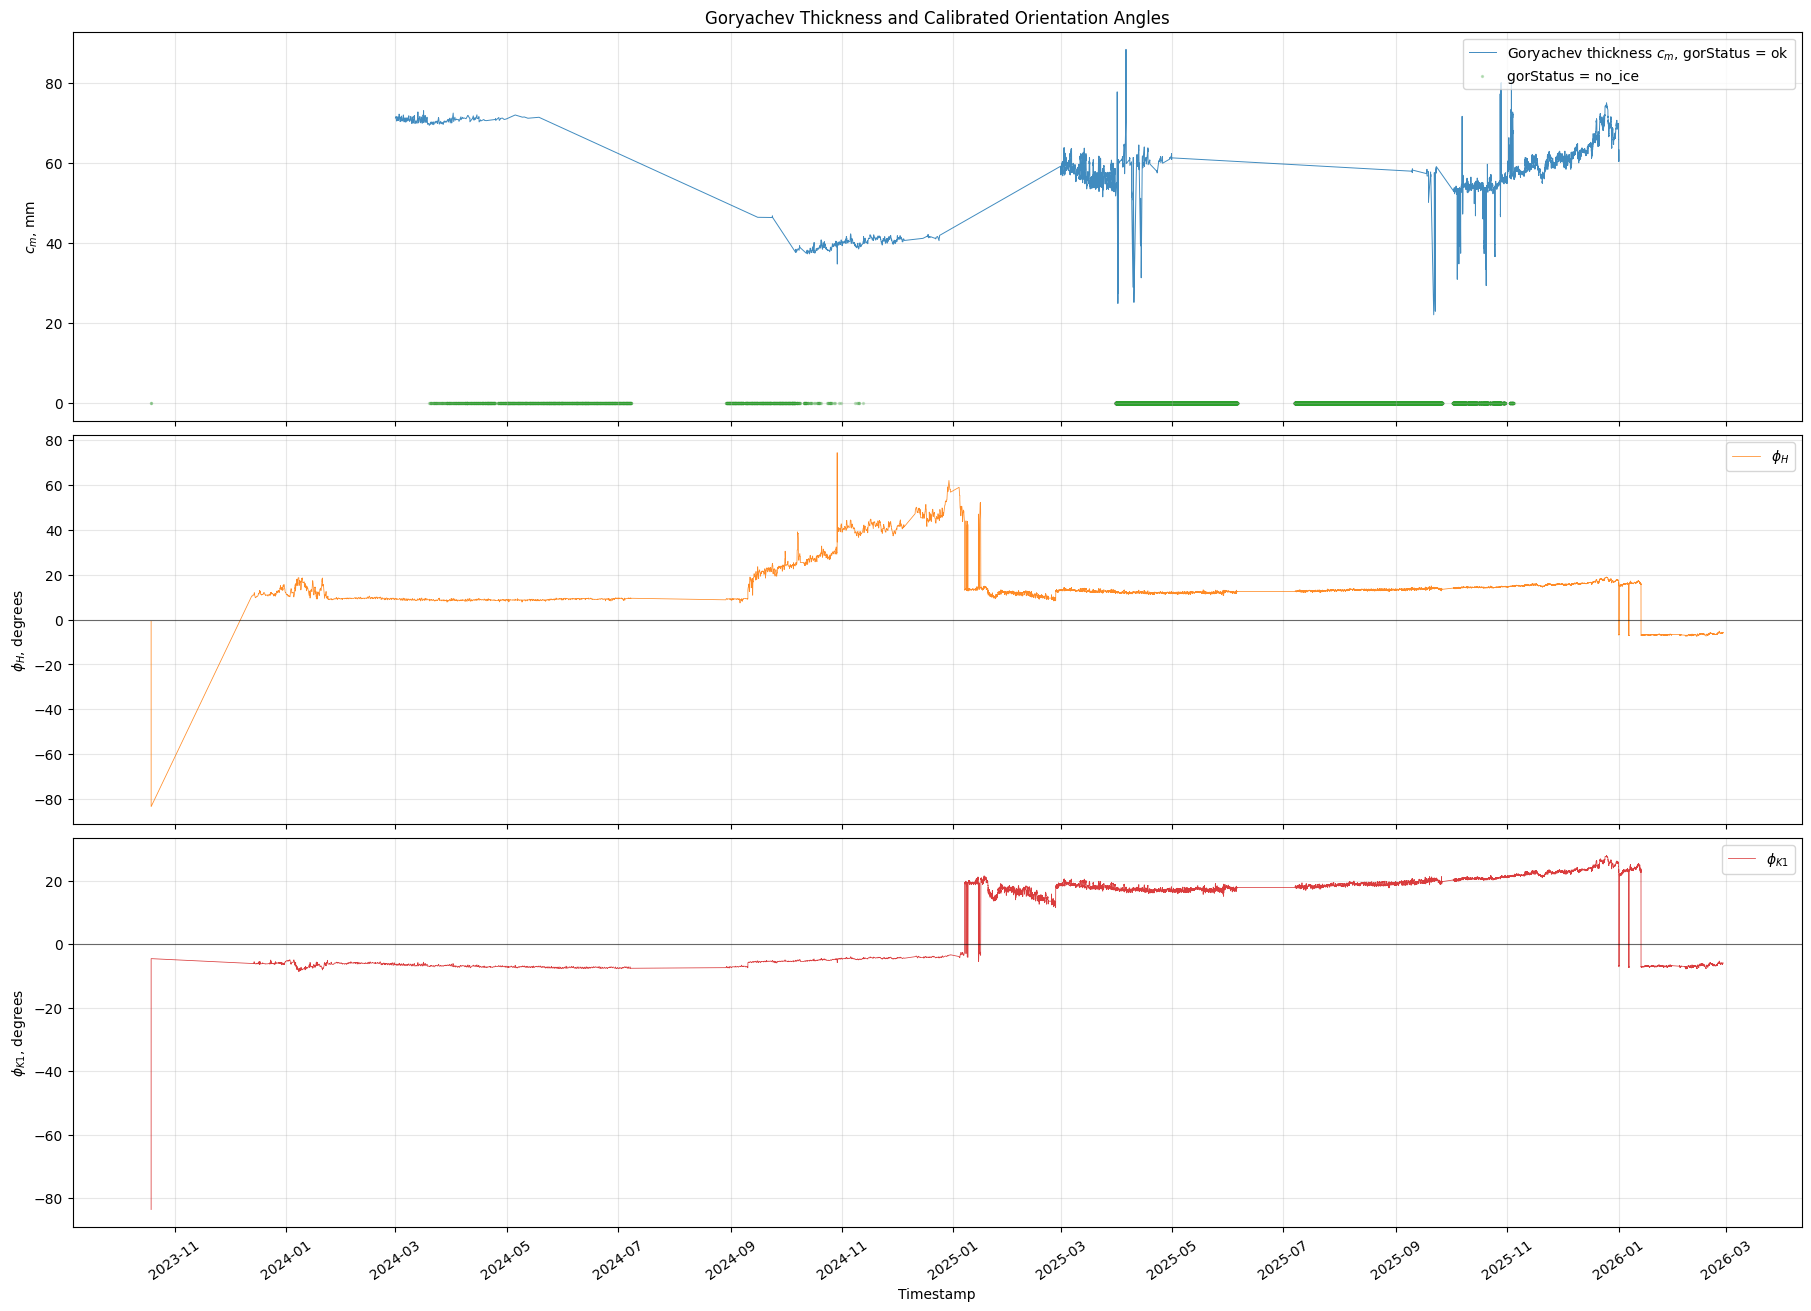

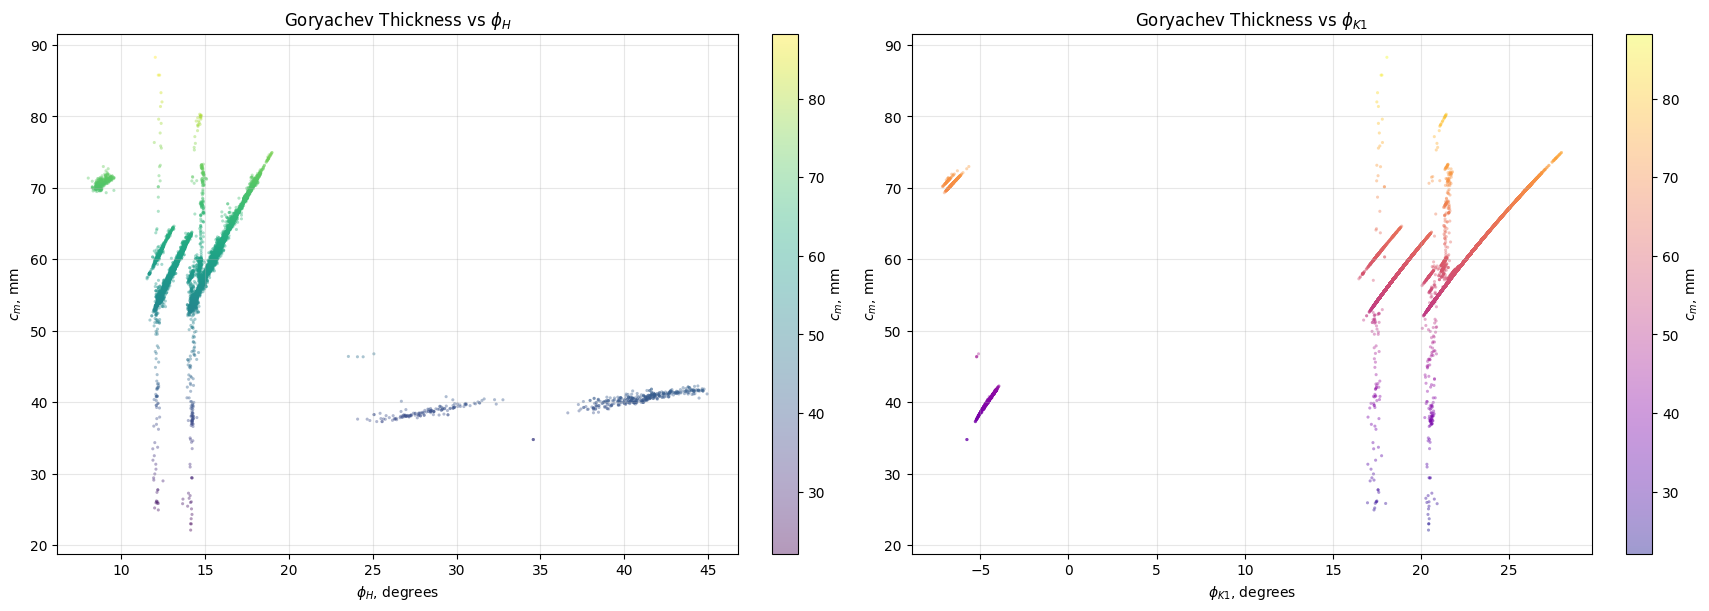

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


# ---------------------------------------------------------------------
# Validate required dataframes.
# ---------------------------------------------------------------------

assert "df_sim" in globals(), (
    "df_sim is not available. "
    "Run the main pipeline first."
)

assert "df_cal" in globals(), (
    "df_cal is not available. "
    "Run the calibration stage / main pipeline first."
)


def resolve_column(
    dataframe: pd.DataFrame,
    candidates: list[str],
    semantic_name: str,
) -> str:
    for column in candidates:
        if column in dataframe.columns:
            return column

    available_candidates = [
        column
        for column in dataframe.columns
        if any(
            token in column.lower()
            for token in [
                "phi",
                "angle",
                "timestamp",
                "gor",
            ]
        )
    ]

    raise KeyError(
        f"Cannot resolve {semantic_name}. "
        f"Expected one of: {candidates}. "
        f"Relevant columns found: "
        f"{available_candidates}"
    )


# ---------------------------------------------------------------------
# Resolve Goryachev columns from df_sim.
# ---------------------------------------------------------------------

SIM_TIMESTAMP_COLUMN = resolve_column(
    dataframe=df_sim,
    candidates=[
        "timestamp",
        "Timestamp",
        "datetime",
    ],
    semantic_name="df_sim timestamp",
)

GOR_CM_COLUMN = resolve_column(
    dataframe=df_sim,
    candidates=[
        "gorCm",
        "goryachevThicknessM",
        "gorCmM",
    ],
    semantic_name="Goryachev thickness",
)

GOR_STATUS_COLUMN = resolve_column(
    dataframe=df_sim,
    candidates=[
        "gorStatus",
        "goryachevStatus",
    ],
    semantic_name="Goryachev status",
)


# ---------------------------------------------------------------------
# Resolve calibrated angle columns from df_cal.
# ---------------------------------------------------------------------

CAL_TIMESTAMP_COLUMN = resolve_column(
    dataframe=df_cal,
    candidates=[
        "timestamp",
        "Timestamp",
        "datetime",
    ],
    semantic_name="df_cal timestamp",
)

PHI_H_COLUMN = resolve_column(
    dataframe=df_cal,
    candidates=[
        "phiHdeg",
        "phiHdeg_cal",
        "phiH_deg",
        "phiH_deg_cal",
    ],
    semantic_name="calibrated phiH angle",
)

PHI_K1_COLUMN = resolve_column(
    dataframe=df_cal,
    candidates=[
        "phiK1deg",
        "phiK1deg_cal",
        "phiK1_deg",
        "phiK1_deg_cal",
    ],
    semantic_name="calibrated phiK1 angle",
)


print("RESOLVED COLUMNS")
print("=" * 72)
print("df_sim timestamp:", SIM_TIMESTAMP_COLUMN)
print("df_sim thickness:", GOR_CM_COLUMN)
print("df_sim status:", GOR_STATUS_COLUMN)
print("df_cal timestamp:", CAL_TIMESTAMP_COLUMN)
print("df_cal phiH:", PHI_H_COLUMN)
print("df_cal phiK1:", PHI_K1_COLUMN)


# ---------------------------------------------------------------------
# Prepare Goryachev simulation output.
# ---------------------------------------------------------------------

df_gor = (
    df_sim[
        [
            SIM_TIMESTAMP_COLUMN,
            GOR_CM_COLUMN,
            GOR_STATUS_COLUMN,
        ]
    ]
    .copy()
    .rename(
        columns={
            SIM_TIMESTAMP_COLUMN: "timestamp",
            GOR_CM_COLUMN: "gorCmM",
            GOR_STATUS_COLUMN: "gorStatus",
        }
    )
)

df_gor["timestamp"] = pd.to_datetime(
    df_gor["timestamp"],
    errors="coerce",
)

df_gor["gorCmM"] = pd.to_numeric(
    df_gor["gorCmM"],
    errors="coerce",
)

df_gor["gorCmMm"] = (
    df_gor["gorCmM"]
    * 1000.0
)

df_gor = (
    df_gor
    .dropna(
        subset=["timestamp"]
    )
    .sort_values("timestamp")
    .reset_index(drop=True)
)


# ---------------------------------------------------------------------
# Prepare calibrated angle data.
# ---------------------------------------------------------------------

df_angles = (
    df_cal[
        [
            CAL_TIMESTAMP_COLUMN,
            PHI_H_COLUMN,
            PHI_K1_COLUMN,
        ]
    ]
    .copy()
    .rename(
        columns={
            CAL_TIMESTAMP_COLUMN: "timestamp",
            PHI_H_COLUMN: "phiHdeg",
            PHI_K1_COLUMN: "phiK1deg",
        }
    )
)

df_angles["timestamp"] = pd.to_datetime(
    df_angles["timestamp"],
    errors="coerce",
)

df_angles["phiHdeg"] = pd.to_numeric(
    df_angles["phiHdeg"],
    errors="coerce",
)

df_angles["phiK1deg"] = pd.to_numeric(
    df_angles["phiK1deg"],
    errors="coerce",
)

df_angles = (
    df_angles
    .dropna(
        subset=["timestamp"]
    )
    .sort_values("timestamp")
    .drop_duplicates(
        subset=["timestamp"],
        keep="last",
    )
    .reset_index(drop=True)
)


# ---------------------------------------------------------------------
# One-to-one merge between simulation output and calibration angles.
# ---------------------------------------------------------------------

assert df_gor["timestamp"].is_unique, (
    "df_sim timestamps are not unique."
)

assert df_angles["timestamp"].is_unique, (
    "df_cal timestamps are not unique."
)


df_gor_plot = (
    df_gor
    .merge(
        df_angles,
        on="timestamp",
        how="left",
        validate="one_to_one",
    )
    .sort_values("timestamp")
    .reset_index(drop=True)
)


n_angle_matched = int(
    df_gor_plot["phiHdeg"]
    .notna()
    .sum()
)

n_angle_unmatched = int(
    df_gor_plot["phiHdeg"]
    .isna()
    .sum()
)

print("\nMERGE AUDIT")
print("=" * 72)
print("df_sim rows:", len(df_gor))
print("df_cal rows:", len(df_angles))
print("Merged rows:", len(df_gor_plot))
print("Rows with phiH match:", n_angle_matched)
print("Rows without phiH match:", n_angle_unmatched)

assert n_angle_unmatched == 0, (
    "Some df_sim rows could not be matched "
    "with calibrated angles."
)


# ---------------------------------------------------------------------
# Status masks.
# ---------------------------------------------------------------------

gor_ok_mask = (
    df_gor_plot["gorStatus"]
    .eq("ok")
    & df_gor_plot["gorCmMm"].notna()
)

gor_no_ice_mask = (
    df_gor_plot["gorStatus"]
    .eq("no_ice")
)

gor_unavailable_mask = (
    ~df_gor_plot["gorStatus"]
    .isin(
        [
            "ok",
            "no_ice",
        ]
    )
)


print("\nGORYACHEV SUMMARY FOR PLOTS")
print("=" * 72)
print("All rows:", len(df_gor_plot))
print("gorStatus = ok:", int(gor_ok_mask.sum()))
print("gorStatus = no_ice:", int(gor_no_ice_mask.sum()))
print(
    "Other Goryachev statuses:",
    int(gor_unavailable_mask.sum()),
)

print(
    "Maximum c_m, mm:",
    round(
        float(
            df_gor_plot.loc[
                gor_ok_mask,
                "gorCmMm",
            ].max()
        ),
        3,
    ),
)


# ---------------------------------------------------------------------
# Figure 1. Thickness and calibrated angles in time.
# ---------------------------------------------------------------------

figure, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(18, 13),
    sharex=True,
    constrained_layout=True,
)


axes[0].plot(
    df_gor_plot.loc[
        gor_ok_mask,
        "timestamp",
    ],
    df_gor_plot.loc[
        gor_ok_mask,
        "gorCmMm",
    ],
    color="tab:blue",
    linewidth=0.70,
    alpha=0.85,
    label=(
        "Goryachev thickness "
        "$c_m$, gorStatus = ok"
    ),
)

axes[0].scatter(
    df_gor_plot.loc[
        gor_no_ice_mask,
        "timestamp",
    ],
    np.zeros(
        int(
            gor_no_ice_mask.sum()
        )
    ),
    color="tab:green",
    s=2,
    alpha=0.25,
    label="gorStatus = no_ice",
)

axes[0].set_title(
    "Goryachev Thickness and Calibrated Orientation Angles"
)

axes[0].set_ylabel(
    "$c_m$, mm"
)

axes[0].grid(
    True,
    alpha=0.30,
)

axes[0].legend(
    loc="upper right",
)


axes[1].plot(
    df_gor_plot["timestamp"],
    df_gor_plot["phiHdeg"],
    color="tab:orange",
    linewidth=0.55,
    alpha=0.90,
    label="$\\phi_H$",
)

axes[1].axhline(
    0.0,
    color="black",
    linewidth=0.8,
    alpha=0.55,
)

axes[1].set_ylabel(
    "$\\phi_H$, degrees"
)

axes[1].grid(
    True,
    alpha=0.30,
)

axes[1].legend(
    loc="upper right",
)


axes[2].plot(
    df_gor_plot["timestamp"],
    df_gor_plot["phiK1deg"],
    color="tab:red",
    linewidth=0.55,
    alpha=0.90,
    label="$\\phi_{K1}$",
)

axes[2].axhline(
    0.0,
    color="black",
    linewidth=0.8,
    alpha=0.55,
)

axes[2].set_ylabel(
    "$\\phi_{K1}$, degrees"
)

axes[2].set_xlabel(
    "Timestamp"
)

axes[2].grid(
    True,
    alpha=0.30,
)

axes[2].legend(
    loc="upper right",
)


axes[2].xaxis.set_major_locator(
    mdates.MonthLocator(
        interval=2,
    )
)

axes[2].xaxis.set_major_formatter(
    mdates.DateFormatter(
        "%Y-%m"
    )
)

for axis in axes:
    axis.tick_params(
        axis="x",
        rotation=35,
    )

plt.show()


# ---------------------------------------------------------------------
# Figure 2. Goryachev thickness vs calibrated angles.
# ---------------------------------------------------------------------

df_gor_scatter = (
    df_gor_plot
    .loc[
        gor_ok_mask
        & df_gor_plot["gorCmMm"].gt(0.0)
    ]
    .dropna(
        subset=[
            "gorCmMm",
            "phiHdeg",
            "phiK1deg",
        ]
    )
    .copy()
)

figure, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(17, 6),
    constrained_layout=True,
)


scatter_phi_h = axes[0].scatter(
    df_gor_scatter["phiHdeg"],
    df_gor_scatter["gorCmMm"],
    c=df_gor_scatter["gorCmMm"],
    cmap="viridis",
    s=5,
    alpha=0.40,
    linewidths=0.0,
)

axes[0].set_title(
    "Goryachev Thickness vs $\\phi_H$"
)

axes[0].set_xlabel(
    "$\\phi_H$, degrees"
)

axes[0].set_ylabel(
    "$c_m$, mm"
)

axes[0].grid(
    True,
    alpha=0.30,
)

figure.colorbar(
    scatter_phi_h,
    ax=axes[0],
    label="$c_m$, mm",
)


scatter_phi_k1 = axes[1].scatter(
    df_gor_scatter["phiK1deg"],
    df_gor_scatter["gorCmMm"],
    c=df_gor_scatter["gorCmMm"],
    cmap="plasma",
    s=5,
    alpha=0.40,
    linewidths=0.0,
)

axes[1].set_title(
    "Goryachev Thickness vs $\\phi_{K1}$"
)

axes[1].set_xlabel(
    "$\\phi_{K1}$, degrees"
)

axes[1].set_ylabel(
    "$c_m$, mm"
)

axes[1].grid(
    True,
    alpha=0.30,
)

figure.colorbar(
    scatter_phi_k1,
    ax=axes[1],
    label="$c_m$, mm",
)

plt.show()

ИНТЕГРАЦИЯ МОДУЛЯ 0042

In [ ]:
import pandas as pd

NO0042_PATH = (
    "/content/"
    "Sensor-VL-module-3-No0042-wide-ffill.csv"
)

df_0042_preview = pd.read_csv(
    NO0042_PATH,
    nrows=20,
)

print(df_0042_preview.columns.tolist())
display(df_0042_preview.head(10))

print(df_0042_preview.dtypes)

['created_at', 'acc', 'boostUP_active', 'e', 'header', 'iideistv', 'iideistva', 'interval', 'iporog', 'ir', 'lsnr', 'noACK', 'rh', 'rssi', 'selfSupply', 'tcab', 'tvozd', 'ugol1', 'ugol2', 'vdd']


,created_at,acc,boostUP_active,e,header,iideistv,iideistva,interval,iporog,ir,lsnr,noACK,rh,rssi,selfSupply,tcab,tvozd,ugol1,ugol2,vdd
0,2023-12-08 06:02:55,28.0,NaN,36.0,6.0,40.0,NaN,3.0,200.0,0.0,-19.5,160.0,76.0,-115.0,1.0,-33.5,-36.0,-3.60,-2.41,3248.0
1,2023-12-08 07:18:06,25.0,NaN,17.0,6.0,43.0,NaN,3.0,200.0,0.0,-19.0,166.0,75.0,-115.0,1.0,-33.9,-36.4,-3.66,-2.41,3312.0
2,2023-12-08 09:10:46,22.0,NaN,18.0,6.0,45.0,NaN,3.0,200.0,0.0,-18.8,175.0,76.0,-115.0,1.0,-33.8,-36.4,-3.72,-2.73,3360.0
3,2023-12-08 14:10:33,22.0,1.0,17.0,6.0,35.0,NaN,3.0,200.0,0.0,-19.0,199.0,76.0,-117.0,1.0,-33.2,-35.7,-3.73,-2.66,3248.0
4,2023-12-09 03:50:18,20.0,0.0,30.0,6.0,39.0,NaN,3.0,200.0,0.0,-16.2,224.0,76.0,-117.0,0.0,-32.0,-34.8,-3.91,-2.55,3232.0
5,2023-12-09 07:22:16,22.0,0.0,19.0,6.0,42.0,NaN,3.0,200.0,0.0,-17.5,241.0,75.0,-117.0,1.0,-32.1,-34.6,-3.80,-2.58,3264.0
6,2023-12-09 07:59:44,21.0,0.0,17.0,6.0,42.0,NaN,3.0,200.0,0.0,-19.0,2.0,75.0,-115.0,1.0,-32.3,-34.7,-3.82,-2.59,3280.0
7,2023-12-09 09:02:11,22.0,0.0,19.0,6.0,42.0,NaN,3.0,200.0,0.0,-18.8,7.0,76.0,-117.0,1.0,-32.0,-34.7,-3.90,-2.73,3312.0
8,2023-12-09 10:42:06,20.0,0.0,18.0,6.0,40.0,NaN,3.0,200.0,0.0,-18.5,7.0,74.0,-117.0,1.0,-32.3,-34.6,-3.84,-2.53,3264.0
9,2023-12-09 11:44:26,21.0,1.0,18.0,6.0,38.0,NaN,3.0,200.0,0.0,-20.0,12.0,73.0,-115.0,1.0,-32.3,-34.7,-3.86,-2.71,3280.0


created_at         object
acc               float64
boostUP_active    float64
e                 float64
header            float64
iideistv          float64
iideistva         float64
interval          float64
iporog            float64
ir                float64
lsnr              float64
noACK             float64
rh                float64
rssi              float64
selfSupply        float64
tcab              float64
tvozd             float64
ugol1             float64
ugol2             float64
vdd               float64
dtype: object


In [ ]:
df_0042_time = pd.read_csv(
    NO0042_PATH,
    usecols=["created_at"],
)

df_0042_time["created_at"] = pd.to_datetime(
    df_0042_time["created_at"],
    errors="coerce",
)

df_0042_time = (
    df_0042_time
    .dropna()
    .sort_values("created_at")
)

dt_minutes = (
    df_0042_time["created_at"]
    .diff()
    .dt.total_seconds()
    / 60.0
)

print(
    dt_minutes.quantile(
        [0.0, 0.01, 0.05, 0.50, 0.95, 0.99, 1.0]
    )
)

0.00        0.000000
0.01        0.000000
0.05        0.000000
0.50        0.133333
0.95      209.233333
0.99      224.623000
1.00    75246.383333
Name: created_at, dtype: float64


In [ ]:
%%writefile /content/hoarfrost_project/src/angle_normalization.py
"""
Angle normalization for Sensor-VL-module-3-No0042.

Safety policy:
- timestamps are deduplicated with keep="last";
- continuity is broken only by configurable long gaps;
- sustained shifts create diagnostic mode candidates;
- only additive offsets are supported;
- sign flips and axis swaps are never applied automatically;
- candidate offsets are applied only when explicitly approved;
- default normalized values equal raw values.

This module is intentionally independent from Goryachev and calibration.
It only prepares raw and optionally approved-normalized ugol1/ugol2.
"""

from __future__ import annotations

from dataclasses import dataclass, field
from typing import Any, Dict, Mapping, Optional

import numpy as np
import pandas as pd


ANGLE_NORMALIZATION_VERSION = "2.0.0"
DEFAULT_SENSOR_ID = "Sensor-VL-module-3-No0042"


@dataclass(frozen=True)
class AngleNormalizationConfig:
    sensor_id: str = DEFAULT_SENSOR_ID
    max_continuity_gap_seconds: float = 6.0 * 3600.0
    sustained_shift_threshold_deg: float = 5.0
    min_sustained_points: int = 4
    local_window_points: int = 3
    transition_merge_seconds: float = 3600.0
    min_mode_points: int = 12
    min_mode_duration_seconds: float = 6.0 * 3600.0
    reference_mode_strategy: str = "first"
    mode: str = "audit_only"
    approved_offsets: Mapping[int, Mapping[str, Any]] = field(
        default_factory=dict
    )


def _coerce_numeric(values: pd.Series) -> pd.Series:
    if pd.api.types.is_numeric_dtype(values):
        return pd.to_numeric(values, errors="coerce")

    prepared = (
        values.astype("string")
        .str.strip()
        .str.replace("\u2212", "-", regex=False)
        .str.replace(",", ".", regex=False)
        .str.replace(r"\s+", "", regex=True)
    )

    return pd.to_numeric(
        prepared,
        errors="coerce",
    )


def _validate_config(
    config: AngleNormalizationConfig,
) -> None:
    allowed_modes = {
        "disabled",
        "audit_only",
        "approved_offsets_only",
    }

    if config.mode not in allowed_modes:
        raise ValueError(
            "Unsupported angle normalization mode: "
            f"{config.mode!r}. "
            f"Allowed modes: {sorted(allowed_modes)}"
        )

    if config.max_continuity_gap_seconds <= 0.0:
        raise ValueError(
            "max_continuity_gap_seconds must be positive."
        )

    if config.sustained_shift_threshold_deg <= 0.0:
        raise ValueError(
            "sustained_shift_threshold_deg must be positive."
        )

    if config.min_sustained_points < 2:
        raise ValueError(
            "min_sustained_points must be at least 2."
        )

    if config.local_window_points < 1:
        raise ValueError(
            "local_window_points must be at least 1."
        )

    if config.reference_mode_strategy not in {
        "first",
        "largest",
    }:
        raise ValueError(
            "reference_mode_strategy must be "
            "'first' or 'largest'."
        )


def prepare_angle_sensor_dataframe(
    dataframe: pd.DataFrame,
    timestamp_column: str = "created_at",
    ugol1_column: str = "ugol1",
    ugol2_column: str = "ugol2",
    sensor_id: str = DEFAULT_SENSOR_ID,
) -> pd.DataFrame:
    required_columns = [
        timestamp_column,
        ugol1_column,
        ugol2_column,
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in dataframe.columns
    ]

    if missing_columns:
        raise KeyError(
            "Angle sensor input is missing columns: "
            f"{missing_columns}. "
            f"Available columns: {list(dataframe.columns)}"
        )

    prepared = (
        dataframe[
            [
                timestamp_column,
                ugol1_column,
                ugol2_column,
            ]
        ]
        .copy()
        .rename(
            columns={
                timestamp_column: "timestamp",
                ugol1_column: "ugol1_raw_deg",
                ugol2_column: "ugol2_raw_deg",
            }
        )
    )

    prepared["timestamp"] = pd.to_datetime(
        prepared["timestamp"],
        errors="coerce",
    )

    prepared["ugol1_raw_deg"] = _coerce_numeric(
        prepared["ugol1_raw_deg"]
    )

    prepared["ugol2_raw_deg"] = _coerce_numeric(
        prepared["ugol2_raw_deg"]
    )

    prepared = (
        prepared
        .dropna(subset=["timestamp"])
        .sort_values("timestamp")
        .drop_duplicates(
            subset=["timestamp"],
            keep="last",
        )
        .reset_index(drop=True)
    )

    prepared["sensor_id"] = str(sensor_id)

    prepared["angles_available"] = (
        prepared["ugol1_raw_deg"].notna()
        & prepared["ugol2_raw_deg"].notna()
    )

    return prepared


def assign_continuous_runs(
    dataframe: pd.DataFrame,
    max_continuity_gap_seconds: float,
) -> pd.DataFrame:
    result = (
        dataframe
        .sort_values("timestamp")
        .reset_index(drop=True)
        .copy()
    )

    gap_seconds = (
        result["timestamp"]
        .diff()
        .dt.total_seconds()
    )

    result["angle_gap_seconds"] = gap_seconds

    result["angle_continuity_break"] = (
        gap_seconds.isna()
        | gap_seconds.gt(
            float(max_continuity_gap_seconds)
        )
        | gap_seconds.le(0.0)
    )

    result["angle_run_id"] = (
        result["angle_continuity_break"]
        .cumsum()
        .astype(int)
    )

    return result


def _detect_shift_candidates_in_run(
    dataframe: pd.DataFrame,
    config: AngleNormalizationConfig,
) -> pd.DataFrame:
    valid = (
        dataframe
        .loc[
            dataframe["angles_available"]
        ]
        .sort_values("timestamp")
        .reset_index(drop=True)
        .copy()
    )

    min_total_points = (
        2 * config.local_window_points
        + config.min_sustained_points
    )

    if len(valid) < min_total_points:
        return pd.DataFrame()

    angle_1 = valid["ugol1_raw_deg"].to_numpy(
        dtype=float
    )

    angle_2 = valid["ugol2_raw_deg"].to_numpy(
        dtype=float
    )

    timestamps = valid["timestamp"].to_numpy()

    records = []

    upper_index = (
        len(valid)
        - config.min_sustained_points
        + 1
    )

    for change_index in range(
        config.local_window_points,
        upper_index,
    ):
        left_slice = slice(
            change_index - config.local_window_points,
            change_index,
        )

        right_slice = slice(
            change_index,
            change_index + config.min_sustained_points,
        )

        left_1 = angle_1[left_slice]
        left_2 = angle_2[left_slice]

        right_1 = angle_1[right_slice]
        right_2 = angle_2[right_slice]

        left_1_median = float(np.median(left_1))
        left_2_median = float(np.median(left_2))

        right_1_median = float(np.median(right_1))
        right_2_median = float(np.median(right_2))

        shift_1 = (
            right_1_median
            - left_1_median
        )

        shift_2 = (
            right_2_median
            - left_2_median
        )

        if (
            abs(shift_1)
            < config.sustained_shift_threshold_deg
            and abs(shift_2)
            < config.sustained_shift_threshold_deg
        ):
            continue

        distance_to_new = np.sqrt(
            (right_1 - right_1_median) ** 2
            + (right_2 - right_2_median) ** 2
        )

        distance_to_old = np.sqrt(
            (right_1 - left_1_median) ** 2
            + (right_2 - left_2_median) ** 2
        )

        consistency = float(
            np.mean(
                distance_to_new
                <= distance_to_old
            )
        )

        if consistency < 0.75:
            continue

        extended_end = min(
            len(valid),
            (
                change_index
                + config.min_sustained_points
                + config.local_window_points
            ),
        )

        extended_1 = angle_1[
            change_index:extended_end
        ]

        extended_2 = angle_2[
            change_index:extended_end
        ]

        extended_distance_to_new = np.sqrt(
            (extended_1 - right_1_median) ** 2
            + (extended_2 - right_2_median) ** 2
        )

        extended_distance_to_old = np.sqrt(
            (extended_1 - left_1_median) ** 2
            + (extended_2 - left_2_median) ** 2
        )

        persistent_fraction = float(
            np.mean(
                extended_distance_to_new
                <= extended_distance_to_old
            )
        )

        if persistent_fraction < 0.75:
            continue

        records.append(
            {
                "angle_run_id": int(
                    valid["angle_run_id"].iloc[0]
                ),
                "change_timestamp": pd.Timestamp(
                    timestamps[change_index]
                ),
                "left_ugol1_median_deg": (
                    left_1_median
                ),
                "left_ugol2_median_deg": (
                    left_2_median
                ),
                "right_ugol1_median_deg": (
                    right_1_median
                ),
                "right_ugol2_median_deg": (
                    right_2_median
                ),
                "shift_ugol1_deg": float(
                    shift_1
                ),
                "shift_ugol2_deg": float(
                    shift_2
                ),
                "shift_vector_norm_deg": float(
                    np.sqrt(
                        shift_1 ** 2
                        + shift_2 ** 2
                    )
                ),
                "level_consistency": consistency,
                "persistent_fraction": (
                    persistent_fraction
                ),
                "candidate_status": (
                    "automatic_candidate_not_approved"
                ),
            }
        )

    return pd.DataFrame(records)


def detect_sustained_shift_candidates(
    dataframe: pd.DataFrame,
    config: AngleNormalizationConfig,
) -> pd.DataFrame:
    candidate_frames = []

    for _, df_run in dataframe.groupby(
        "angle_run_id",
        sort=True,
    ):
        candidates = _detect_shift_candidates_in_run(
            dataframe=df_run,
            config=config,
        )

        if not candidates.empty:
            candidate_frames.append(candidates)

    if not candidate_frames:
        return pd.DataFrame(
            columns=[
                "angle_run_id",
                "change_timestamp",
                "left_ugol1_median_deg",
                "left_ugol2_median_deg",
                "right_ugol1_median_deg",
                "right_ugol2_median_deg",
                "shift_ugol1_deg",
                "shift_ugol2_deg",
                "shift_vector_norm_deg",
                "level_consistency",
                "persistent_fraction",
                "candidate_status",
            ]
        )

    raw_candidates = (
        pd.concat(
            candidate_frames,
            ignore_index=True,
        )
        .sort_values(
            [
                "angle_run_id",
                "change_timestamp",
            ]
        )
        .reset_index(drop=True)
    )

    kept_rows = []

    for run_id, df_run in raw_candidates.groupby(
        "angle_run_id",
        sort=True,
    ):
        previous_timestamp: Optional[pd.Timestamp] = None

        for _, row in df_run.iterrows():
            timestamp = pd.Timestamp(
                row["change_timestamp"]
            )

            if (
                previous_timestamp is not None
                and (
                    timestamp - previous_timestamp
                ).total_seconds()
                <= config.transition_merge_seconds
            ):
                continue

            kept_rows.append(row.to_dict())
            previous_timestamp = timestamp

    return (
        pd.DataFrame(kept_rows)
        .sort_values(
            [
                "angle_run_id",
                "change_timestamp",
            ]
        )
        .reset_index(drop=True)
        if kept_rows
        else raw_candidates.iloc[0:0].copy()
    )


def build_angle_modes(
    dataframe: pd.DataFrame,
    shift_candidates: pd.DataFrame,
    config: AngleNormalizationConfig,
) -> pd.DataFrame:
    records = []
    next_mode_id = 0

    candidate_times_by_run: Dict[
        int,
        list[pd.Timestamp],
    ] = {}

    if not shift_candidates.empty:
        for run_id, df_run in shift_candidates.groupby(
            "angle_run_id",
            sort=True,
        ):
            candidate_times_by_run[int(run_id)] = [
                pd.Timestamp(value)
                for value in df_run[
                    "change_timestamp"
                ].tolist()
            ]

    for run_id, df_run in dataframe.groupby(
        "angle_run_id",
        sort=True,
    ):
        df_run = (
            df_run
            .sort_values("timestamp")
            .reset_index(drop=True)
        )

        change_times = candidate_times_by_run.get(
            int(run_id),
            [],
        )

        mode_start = pd.Timestamp(
            df_run["timestamp"].min()
        )

        for change_time in change_times:
            df_mode = df_run.loc[
                (
                    df_run["timestamp"]
                    >= mode_start
                )
                & (
                    df_run["timestamp"]
                    < change_time
                )
            ]

            if not df_mode.empty:
                records.append(
                    {
                        "angle_mode_id": next_mode_id,
                        "angle_run_id": int(run_id),
                        "mode_start": df_mode[
                            "timestamp"
                        ].min(),
                        "mode_end": df_mode[
                            "timestamp"
                        ].max(),
                        "mode_length_points": int(
                            len(df_mode)
                        ),
                    }
                )

                next_mode_id += 1

            mode_start = pd.Timestamp(change_time)

        df_last = df_run.loc[
            df_run["timestamp"]
            >= mode_start
        ]

        if not df_last.empty:
            records.append(
                {
                    "angle_mode_id": next_mode_id,
                    "angle_run_id": int(run_id),
                    "mode_start": df_last[
                        "timestamp"
                    ].min(),
                    "mode_end": df_last[
                        "timestamp"
                    ].max(),
                    "mode_length_points": int(
                        len(df_last)
                    ),
                }
            )

            next_mode_id += 1

    modes = pd.DataFrame(records)

    if modes.empty:
        return pd.DataFrame(
            columns=[
                "angle_mode_id",
                "angle_run_id",
                "mode_start",
                "mode_end",
                "mode_length_points",
                "mode_duration_seconds",
                "mode_is_long_enough",
                "reference_mode_id",
            ]
        )

    modes["mode_duration_seconds"] = (
        modes["mode_end"]
        - modes["mode_start"]
    ).dt.total_seconds()

    modes["mode_is_long_enough"] = (
        modes["mode_length_points"].ge(
            config.min_mode_points
        )
        & modes["mode_duration_seconds"].ge(
            config.min_mode_duration_seconds
        )
    )

    eligible_modes = modes.loc[
        modes["mode_is_long_enough"]
    ].copy()

    if eligible_modes.empty:
        reference_mode_id = int(
            modes["angle_mode_id"].iloc[0]
        )

    elif config.reference_mode_strategy == "largest":
        reference_mode_id = int(
            eligible_modes.loc[
                eligible_modes[
                    "mode_length_points"
                ].idxmax(),
                "angle_mode_id",
            ]
        )

    else:
        reference_mode_id = int(
            eligible_modes[
                "angle_mode_id"
            ].min()
        )

    modes["reference_mode_id"] = reference_mode_id

    return modes


def assign_modes_to_rows(
    dataframe: pd.DataFrame,
    modes: pd.DataFrame,
) -> pd.DataFrame:
    result = dataframe.copy()

    result["angle_mode_id"] = pd.Series(
        pd.NA,
        index=result.index,
        dtype="Int64",
    )

    for _, mode in modes.iterrows():
        mask = (
            result["angle_run_id"].eq(
                int(mode["angle_run_id"])
            )
            & result["timestamp"].ge(
                pd.Timestamp(
                    mode["mode_start"]
                )
            )
            & result["timestamp"].le(
                pd.Timestamp(
                    mode["mode_end"]
                )
            )
        )

        result.loc[
            mask,
            "angle_mode_id",
        ] = int(mode["angle_mode_id"])

    return result


def estimate_offset_candidates(
    dataframe: pd.DataFrame,
    modes: pd.DataFrame,
) -> pd.DataFrame:
    if dataframe.empty or modes.empty:
        return pd.DataFrame()

    reference_mode_id = int(
        modes["reference_mode_id"].iloc[0]
    )

    reference_rows = dataframe.loc[
        dataframe["angle_mode_id"].eq(
            reference_mode_id
        )
        & dataframe["angles_available"]
    ]

    if reference_rows.empty:
        return pd.DataFrame()

    reference_ugol1 = float(
        reference_rows["ugol1_raw_deg"].median()
    )

    reference_ugol2 = float(
        reference_rows["ugol2_raw_deg"].median()
    )

    records = []

    for _, mode in modes.iterrows():
        mode_id = int(mode["angle_mode_id"])

        mode_rows = dataframe.loc[
            dataframe["angle_mode_id"].eq(
                mode_id
            )
            & dataframe["angles_available"]
        ]

        if mode_rows.empty:
            continue

        mode_ugol1 = float(
            mode_rows["ugol1_raw_deg"].median()
        )

        mode_ugol2 = float(
            mode_rows["ugol2_raw_deg"].median()
        )

        offset_ugol1 = (
            mode_ugol1
            - reference_ugol1
        )

        offset_ugol2 = (
            mode_ugol2
            - reference_ugol2
        )

        records.append(
            {
                "angle_mode_id": mode_id,
                "reference_mode_id": (
                    reference_mode_id
                ),
                "candidate_transform": "offset",
                "candidate_offset_ugol1_deg": (
                    float(offset_ugol1)
                ),
                "candidate_offset_ugol2_deg": (
                    float(offset_ugol2)
                ),
                "candidate_offset_norm_deg": float(
                    np.sqrt(
                        offset_ugol1 ** 2
                        + offset_ugol2 ** 2
                    )
                ),
                "candidate_status": (
                    "automatic_candidate_not_approved"
                ),
            }
        )

    return pd.DataFrame(records)


def _approved_offset_for_mode(
    mode_id: int,
    config: AngleNormalizationConfig,
) -> Optional[Mapping[str, Any]]:
    specification = config.approved_offsets.get(
        int(mode_id)
    )

    if not specification:
        return None

    if not bool(
        specification.get(
            "approved",
            False,
        )
    ):
        return None

    if specification.get(
        "transform",
        "offset",
    ) != "offset":
        raise ValueError(
            "Only approved additive offset "
            "transforms are supported."
        )

    return specification


def apply_approved_offsets(
    dataframe: pd.DataFrame,
    config: AngleNormalizationConfig,
) -> pd.DataFrame:
    result = dataframe.copy()

    result["ugol1_norm_deg"] = result[
        "ugol1_raw_deg"
    ]

    result["ugol2_norm_deg"] = result[
        "ugol2_raw_deg"
    ]

    result["angle_transform"] = "identity"

    result["angle_offset_ugol1_deg"] = 0.0
    result["angle_offset_ugol2_deg"] = 0.0

    result["angle_normalization_approved"] = False

    if config.mode != "approved_offsets_only":
        result["angle_normalization_quality"] = (
            "raw_or_audit_only"
        )
        return result

    for mode_id in (
        result["angle_mode_id"]
        .dropna()
        .astype(int)
        .unique()
    ):
        specification = _approved_offset_for_mode(
            mode_id=int(mode_id),
            config=config,
        )

        if specification is None:
            continue

        offset_ugol1 = float(
            specification.get(
                "offset_ugol1_deg",
                0.0,
            )
        )

        offset_ugol2 = float(
            specification.get(
                "offset_ugol2_deg",
                0.0,
            )
        )

        mask = result["angle_mode_id"].eq(
            int(mode_id)
        )

        result.loc[
            mask,
            "ugol1_norm_deg",
        ] = (
            result.loc[
                mask,
                "ugol1_raw_deg",
            ]
            - offset_ugol1
        )

        result.loc[
            mask,
            "ugol2_norm_deg",
        ] = (
            result.loc[
                mask,
                "ugol2_raw_deg",
            ]
            - offset_ugol2
        )

        result.loc[
            mask,
            "angle_transform",
        ] = "approved_offset"

        result.loc[
            mask,
            "angle_offset_ugol1_deg",
        ] = offset_ugol1

        result.loc[
            mask,
            "angle_offset_ugol2_deg",
        ] = offset_ugol2

        result.loc[
            mask,
            "angle_normalization_approved",
        ] = True

    result["angle_normalization_quality"] = np.where(
        result["angle_normalization_approved"],
        "approved_offset",
        "raw_pending_approval",
    )

    return result


def normalize_sensor_angles(
    dataframe: pd.DataFrame,
    config: AngleNormalizationConfig = (
        AngleNormalizationConfig()
    ),
    timestamp_column: str = "created_at",
    ugol1_column: str = "ugol1",
    ugol2_column: str = "ugol2",
) -> Dict[str, Any]:
    _validate_config(config)

    prepared = prepare_angle_sensor_dataframe(
        dataframe=dataframe,
        timestamp_column=timestamp_column,
        ugol1_column=ugol1_column,
        ugol2_column=ugol2_column,
        sensor_id=config.sensor_id,
    )

    prepared = assign_continuous_runs(
        dataframe=prepared,
        max_continuity_gap_seconds=(
            config.max_continuity_gap_seconds
        ),
    )

    if config.mode == "disabled":
        prepared["angle_mode_id"] = pd.Series(
            0,
            index=prepared.index,
            dtype="Int64",
        )

        prepared["reference_mode_id"] = 0

        prepared["ugol1_norm_deg"] = prepared[
            "ugol1_raw_deg"
        ]

        prepared["ugol2_norm_deg"] = prepared[
            "ugol2_raw_deg"
        ]

        prepared["angle_transform"] = "disabled"

        prepared["angle_offset_ugol1_deg"] = 0.0
        prepared["angle_offset_ugol2_deg"] = 0.0

        prepared["angle_normalization_approved"] = False

        prepared["angle_normalization_quality"] = (
            "normalization_disabled"
        )

        return {
            "normalized": prepared,
            "shift_candidates": pd.DataFrame(),
            "modes": pd.DataFrame(),
            "offset_candidates": pd.DataFrame(),
            "summary": {
                "angle_normalization_version": (
                    ANGLE_NORMALIZATION_VERSION
                ),
                "mode": config.mode,
                "sensor_id": config.sensor_id,
                "n_input_rows": int(len(dataframe)),
                "n_output_rows": int(len(prepared)),
                "n_runs": int(
                    prepared["angle_run_id"]
                    .nunique()
                ),
                "n_shift_candidates": 0,
                "n_modes": 0,
                "n_approved_offset_rows": 0,
            },
        }

    shift_candidates = detect_sustained_shift_candidates(
        dataframe=prepared,
        config=config,
    )

    modes = build_angle_modes(
        dataframe=prepared,
        shift_candidates=shift_candidates,
        config=config,
    )

    with_modes = assign_modes_to_rows(
        dataframe=prepared,
        modes=modes,
    )

    if modes.empty:
        with_modes["reference_mode_id"] = pd.Series(
            pd.NA,
            index=with_modes.index,
            dtype="Int64",
        )
    else:
        with_modes["reference_mode_id"] = int(
            modes["reference_mode_id"].iloc[0]
        )

    offset_candidates = estimate_offset_candidates(
        dataframe=with_modes,
        modes=modes,
    )

    normalized = apply_approved_offsets(
        dataframe=with_modes,
        config=config,
    )

    summary = {
        "angle_normalization_version": (
            ANGLE_NORMALIZATION_VERSION
        ),
        "mode": config.mode,
        "sensor_id": config.sensor_id,
        "n_input_rows": int(len(dataframe)),
        "n_output_rows": int(len(normalized)),
        "n_angles_available_rows": int(
            normalized["angles_available"].sum()
        ),
        "n_runs": int(
            normalized["angle_run_id"].nunique()
        ),
        "n_shift_candidates": int(
            len(shift_candidates)
        ),
        "n_modes": int(len(modes)),
        "n_approved_offset_rows": int(
            normalized[
                "angle_normalization_approved"
            ].sum()
        ),
    }

    return {
        "normalized": normalized,
        "shift_candidates": shift_candidates,
        "modes": modes,
        "offset_candidates": offset_candidates,
        "summary": summary,
    }

Writing /content/hoarfrost_project/src/angle_normalization.py


In [ ]:
import importlib
import sys


for module_name in list(sys.modules):
    if (
        module_name == "src.angle_normalization"
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()

from src.angle_normalization import (
    ANGLE_NORMALIZATION_VERSION,
    AngleNormalizationConfig,
    normalize_sensor_angles,
)

print(
    "Angle normalization import passed."
)

print(
    "Module version:",
    ANGLE_NORMALIZATION_VERSION,
)

Angle normalization import passed.
Module version: 2.0.0


In [ ]:
from pathlib import Path

import pandas as pd


SENSOR_0042_CSV_PATH = Path(
    "/content/"
    "Sensor-VL-module-3-No0042-wide-ffill.csv"
)

assert SENSOR_0042_CSV_PATH.exists(), (
    "No0042 CSV was not found: "
    f"{SENSOR_0042_CSV_PATH}"
)


df_0042_raw = pd.read_csv(
    SENSOR_0042_CSV_PATH,
    low_memory=False,
)


angle_0042_config = AngleNormalizationConfig(
    sensor_id="Sensor-VL-module-3-No0042",
    max_continuity_gap_seconds=6.0 * 3600.0,
    sustained_shift_threshold_deg=5.0,
    min_sustained_points=4,
    local_window_points=3,
    transition_merge_seconds=3600.0,
    min_mode_points=12,
    min_mode_duration_seconds=6.0 * 3600.0,
    reference_mode_strategy="first",
    mode="audit_only",
    approved_offsets={},
)


angle_0042_result = normalize_sensor_angles(
    dataframe=df_0042_raw,
    config=angle_0042_config,
    timestamp_column="created_at",
    ugol1_column="ugol1",
    ugol2_column="ugol2",
)


df_0042_normalized = angle_0042_result[
    "normalized"
]

df_0042_shift_candidates = angle_0042_result[
    "shift_candidates"
]

df_0042_modes = angle_0042_result[
    "modes"
]

df_0042_offset_candidates = angle_0042_result[
    "offset_candidates"
]

angle_0042_summary = angle_0042_result[
    "summary"
]


print("ANGLE 0042 NORMALIZATION SUMMARY")
print("=" * 78)

for key, value in angle_0042_summary.items():
    print(f"{key}: {value}")


print("\nNORMALIZED 0042 PREVIEW")
display(
    df_0042_normalized.head(10)
)


print("\nMODE PREVIEW")
display(
    df_0042_modes.head(20)
)


print("\nSHIFT-CANDIDATE PREVIEW")
display(
    df_0042_shift_candidates.head(20)
)


print("\nOFFSET-CANDIDATE PREVIEW")
display(
    df_0042_offset_candidates.head(20)
)


assert (
    df_0042_normalized["timestamp"]
    .is_monotonic_increasing
)

assert (
    df_0042_normalized["timestamp"]
    .is_unique
)

assert (
    np.allclose(
        df_0042_normalized["ugol1_raw_deg"],
        df_0042_normalized["ugol1_norm_deg"],
        equal_nan=True,
    )
)

assert (
    np.allclose(
        df_0042_normalized["ugol2_raw_deg"],
        df_0042_normalized["ugol2_norm_deg"],
        equal_nan=True,
    )
)

assert not bool(
    df_0042_normalized[
        "angle_normalization_approved"
    ].any()
)

print(
    "\nAudit-only safety checks passed: "
    "no offset was automatically applied."
)

ANGLE 0042 NORMALIZATION SUMMARY
angle_normalization_version: 2.0.0
mode: audit_only
sensor_id: Sensor-VL-module-3-No0042
n_input_rows: 31665
n_output_rows: 20332
n_angles_available_rows: 20331
n_runs: 150
n_shift_candidates: 34
n_modes: 184
n_approved_offset_rows: 0

NORMALIZED 0042 PREVIEW


,timestamp,ugol1_raw_deg,ugol2_raw_deg,sensor_id,angles_available,angle_gap_seconds,angle_continuity_break,angle_run_id,angle_mode_id,reference_mode_id,ugol1_norm_deg,ugol2_norm_deg,angle_transform,angle_offset_ugol1_deg,angle_offset_ugol2_deg,angle_normalization_approved,angle_normalization_quality
0,2023-12-08 06:02:55,-3.60,-2.41,Sensor-VL-module-3-No0042,True,NaN,True,1,0,2,-3.60,-2.41,identity,0.0,0.0,False,raw_or_audit_only
1,2023-12-08 07:18:06,-3.66,-2.41,Sensor-VL-module-3-No0042,True,4511.0,False,1,0,2,-3.66,-2.41,identity,0.0,0.0,False,raw_or_audit_only
2,2023-12-08 09:10:46,-3.72,-2.73,Sensor-VL-module-3-No0042,True,6760.0,False,1,0,2,-3.72,-2.73,identity,0.0,0.0,False,raw_or_audit_only
3,2023-12-08 14:10:33,-3.73,-2.66,Sensor-VL-module-3-No0042,True,17987.0,False,1,0,2,-3.73,-2.66,identity,0.0,0.0,False,raw_or_audit_only
4,2023-12-09 03:50:18,-3.91,-2.55,Sensor-VL-module-3-No0042,True,49185.0,True,2,1,2,-3.91,-2.55,identity,0.0,0.0,False,raw_or_audit_only
5,2023-12-09 07:22:16,-3.80,-2.58,Sensor-VL-module-3-No0042,True,12718.0,False,2,1,2,-3.80,-2.58,identity,0.0,0.0,False,raw_or_audit_only
6,2023-12-09 07:59:44,-3.82,-2.59,Sensor-VL-module-3-No0042,True,2248.0,False,2,1,2,-3.82,-2.59,identity,0.0,0.0,False,raw_or_audit_only
7,2023-12-09 09:02:11,-3.90,-2.73,Sensor-VL-module-3-No0042,True,3747.0,False,2,1,2,-3.90,-2.73,identity,0.0,0.0,False,raw_or_audit_only
8,2023-12-09 10:42:06,-3.84,-2.53,Sensor-VL-module-3-No0042,True,5995.0,False,2,1,2,-3.84,-2.53,identity,0.0,0.0,False,raw_or_audit_only
9,2023-12-09 11:44:26,-3.86,-2.71,Sensor-VL-module-3-No0042,True,3740.0,False,2,1,2,-3.86,-2.71,identity,0.0,0.0,False,raw_or_audit_only



MODE PREVIEW


,angle_mode_id,angle_run_id,mode_start,mode_end,mode_length_points,mode_duration_seconds,mode_is_long_enough,reference_mode_id
0,0,1,2023-12-08 06:02:55,2023-12-08 14:10:33,4,29258.0,False,2
1,1,2,2023-12-09 03:50:18,2023-12-09 15:29:05,8,41927.0,False,2
2,2,3,2023-12-10 21:57:55,2023-12-11 10:24:16,12,44781.0,True,2
3,3,4,2023-12-12 20:04:26,2023-12-12 20:04:26,1,0.0,False,2
4,4,5,2023-12-13 07:09:23,2023-12-14 16:27:41,10,119898.0,False,2
5,5,6,2023-12-14 23:54:15,2023-12-25 14:10:52,241,915397.0,True,2
6,6,7,2023-12-25 21:35:06,2023-12-28 22:05:20,54,261014.0,True,2
7,7,8,2023-12-29 05:42:38,2023-12-29 17:04:48,5,40930.0,False,2
8,8,9,2023-12-30 00:39:33,2023-12-30 12:00:34,4,40861.0,False,2
9,9,10,2023-12-30 19:37:20,2023-12-30 19:37:21,2,1.0,False,2



SHIFT-CANDIDATE PREVIEW


,angle_run_id,change_timestamp,left_ugol1_median_deg,left_ugol2_median_deg,right_ugol1_median_deg,right_ugol2_median_deg,shift_ugol1_deg,shift_ugol2_deg,shift_vector_norm_deg,level_consistency,persistent_fraction,candidate_status
0,90,2025-01-07 04:14:48,-4.47,-5.10,9.340,-8.100,13.810,-3.000,14.132095,0.75,0.857143,automatic_candidate_not_approved
1,90,2025-01-07 05:16:00,-4.47,-5.10,9.340,-8.100,13.810,-3.000,14.132095,1.00,1.000000,automatic_candidate_not_approved
2,90,2025-01-09 02:44:34,10.40,-8.80,-4.490,-6.220,-14.890,2.580,15.111866,0.75,0.857143,automatic_candidate_not_approved
3,90,2025-01-09 06:34:10,10.39,-8.80,-4.405,-6.220,-14.795,2.580,15.018270,1.00,1.000000,automatic_candidate_not_approved
4,93,2025-01-17 02:59:49,-4.63,-7.12,10.710,-9.025,15.340,-1.905,15.457834,1.00,1.000000,automatic_candidate_not_approved
5,93,2025-01-17 11:01:59,10.62,-8.95,-4.210,-6.525,-14.830,2.425,15.026960,0.75,0.857143,automatic_candidate_not_approved
6,93,2025-01-17 14:54:41,10.62,-8.98,-4.140,-6.990,-14.760,1.990,14.893546,1.00,1.000000,automatic_candidate_not_approved
7,94,2025-01-19 07:59:17,10.72,-9.03,-4.395,-7.220,-15.115,1.810,15.222987,0.75,0.857143,automatic_candidate_not_approved
8,94,2025-01-19 23:08:30,-4.36,-7.20,10.630,-8.975,14.990,-1.775,15.094725,0.75,0.857143,automatic_candidate_not_approved
9,94,2025-01-20 02:12:04,-4.43,-7.24,10.640,-9.005,15.070,-1.765,15.173006,1.00,1.000000,automatic_candidate_not_approved



OFFSET-CANDIDATE PREVIEW


,angle_mode_id,reference_mode_id,candidate_transform,candidate_offset_ugol1_deg,candidate_offset_ugol2_deg,candidate_offset_norm_deg,candidate_status
0,0,2,offset,0.125,0.010,0.125399,automatic_candidate_not_approved
1,1,2,offset,-0.050,-0.050,0.070711,automatic_candidate_not_approved
2,2,2,offset,0.000,0.000,0.000000,automatic_candidate_not_approved
3,3,2,offset,-0.315,-0.805,0.864436,automatic_candidate_not_approved
4,4,2,offset,-0.415,-0.735,0.844068,automatic_candidate_not_approved
5,5,2,offset,-1.515,-2.065,2.561142,automatic_candidate_not_approved
6,6,2,offset,-1.200,-2.325,2.616415,automatic_candidate_not_approved
7,7,2,offset,-0.835,-2.615,2.745077,automatic_candidate_not_approved
8,8,2,offset,-0.665,-2.285,2.379800,automatic_candidate_not_approved
9,9,2,offset,-0.165,-2.995,2.999542,automatic_candidate_not_approved



Audit-only safety checks passed: no offset was automatically applied.


In [ ]:
%%writefile -a /content/hoarfrost_project/src/data_normalization.py


# ---------------------------------------------------------------------------
# Optional Sensor No0042 normalized-angle integration.
#
# Added after the frozen legacy normalization/METAR/solar builders.
# Default behavior is fully disabled and preserves the legacy No0039 path.
# ---------------------------------------------------------------------------

from dataclasses import field as _angle0042_field
from typing import Mapping as _Angle0042Mapping


ANGLE_0042_INTEGRATION_VERSION = "1.0.0"
ANGLE_0042_DEFAULT_MAX_AGE_SECONDS = 3 * 60 * 60


@dataclass(frozen=True)
class Angle0042IntegrationConfig:
    enabled: bool = False
    use_normalized_0042_as_active_angles: bool = False
    max_angle_age_seconds: float = (
        ANGLE_0042_DEFAULT_MAX_AGE_SECONDS
    )
    normalization_mode: str = "audit_only"
    max_continuity_gap_seconds: float = 6.0 * 3600.0
    sustained_shift_threshold_deg: float = 5.0
    min_sustained_points: int = 4
    local_window_points: int = 3
    transition_merge_seconds: float = 3600.0
    min_mode_points: int = 12
    min_mode_duration_seconds: float = 6.0 * 3600.0
    reference_mode_strategy: str = "first"
    approved_offsets: _Angle0042Mapping[
        int,
        _Angle0042Mapping[str, Any],
    ] = _angle0042_field(
        default_factory=dict
    )


def _angle0042_normalization_config(
    config: Angle0042IntegrationConfig,
) -> Any:
    from src.angle_normalization import (
        AngleNormalizationConfig,
    )

    return AngleNormalizationConfig(
        sensor_id="Sensor-VL-module-3-No0042",
        max_continuity_gap_seconds=float(
            config.max_continuity_gap_seconds
        ),
        sustained_shift_threshold_deg=float(
            config.sustained_shift_threshold_deg
        ),
        min_sustained_points=int(
            config.min_sustained_points
        ),
        local_window_points=int(
            config.local_window_points
        ),
        transition_merge_seconds=float(
            config.transition_merge_seconds
        ),
        min_mode_points=int(
            config.min_mode_points
        ),
        min_mode_duration_seconds=float(
            config.min_mode_duration_seconds
        ),
        reference_mode_strategy=str(
            config.reference_mode_strategy
        ),
        mode=str(
            config.normalization_mode
        ),
        approved_offsets=dict(
            config.approved_offsets
        ),
    )


def _validate_angle0042_integration_config(
    config: Angle0042IntegrationConfig,
) -> None:
    if config.max_angle_age_seconds <= 0.0:
        raise ValueError(
            "max_angle_age_seconds must be positive."
        )

    allowed_modes = {
        "disabled",
        "audit_only",
        "approved_offsets_only",
    }

    if config.normalization_mode not in allowed_modes:
        raise ValueError(
            "Unsupported No0042 normalization mode: "
            f"{config.normalization_mode!r}."
        )

    if (
        config.use_normalized_0042_as_active_angles
        and not config.enabled
    ):
        raise ValueError(
            "No0042 active-angle substitution requires "
            "enabled=True."
        )

    if (
        config.use_normalized_0042_as_active_angles
        and config.normalization_mode
        != "approved_offsets_only"
    ):
        raise ValueError(
            "Active No0042 substitution is permitted only "
            "when normalization_mode="
            "'approved_offsets_only'."
        )


def _prepare_no0042_angle_table(
    sensor_angle_0042_csv_path: str | Path,
    config: Angle0042IntegrationConfig,
) -> tuple[
    pd.DataFrame,
    pd.DataFrame,
    pd.DataFrame,
    pd.DataFrame,
    Dict[str, Any],
]:
    from src.angle_normalization import (
        normalize_sensor_angles,
    )

    raw_0042 = read_csv_auto(
        sensor_angle_0042_csv_path
    )

    normalized_result = normalize_sensor_angles(
        dataframe=raw_0042,
        config=_angle0042_normalization_config(
            config
        ),
        timestamp_column="created_at",
        ugol1_column="ugol1",
        ugol2_column="ugol2",
    )

    normalized = normalized_result[
        "normalized"
    ].copy()

    normalized["angle0042Timestamp"] = pd.to_datetime(
        normalized["timestamp"],
        errors="coerce",
    )

    normalized = (
        normalized
        .dropna(
            subset=["angle0042Timestamp"]
        )
        .sort_values("angle0042Timestamp")
        .drop_duplicates(
            subset=["angle0042Timestamp"],
            keep="last",
        )
        .reset_index(drop=True)
    )

    normalized = normalized.rename(
        columns={
            "ugol1_raw_deg": (
                "ugol1DegRaw0042"
            ),
            "ugol2_raw_deg": (
                "ugol2DegRaw0042"
            ),
            "ugol1_norm_deg": (
                "ugol1DegNorm0042"
            ),
            "ugol2_norm_deg": (
                "ugol2DegNorm0042"
            ),
            "angle_run_id": (
                "angle0042RunId"
            ),
            "angle_mode_id": (
                "angle0042ModeId"
            ),
            "reference_mode_id": (
                "angle0042ReferenceModeId"
            ),
            "angle_transform": (
                "angle0042Transform"
            ),
            "angle_offset_ugol1_deg": (
                "angle0042OffsetUgol1Deg"
            ),
            "angle_offset_ugol2_deg": (
                "angle0042OffsetUgol2Deg"
            ),
            "angle_normalization_approved": (
                "angle0042NormalizationApproved"
            ),
            "angle_normalization_quality": (
                "angle0042NormalizationQuality"
            ),
        }
    )

    selected_columns = [
        "angle0042Timestamp",
        "ugol1DegRaw0042",
        "ugol2DegRaw0042",
        "ugol1DegNorm0042",
        "ugol2DegNorm0042",
        "angles_available",
        "angle_gap_seconds",
        "angle_continuity_break",
        "angle0042RunId",
        "angle0042ModeId",
        "angle0042ReferenceModeId",
        "angle0042Transform",
        "angle0042OffsetUgol1Deg",
        "angle0042OffsetUgol2Deg",
        "angle0042NormalizationApproved",
        "angle0042NormalizationQuality",
    ]

    selected_columns = [
        column
        for column in selected_columns
        if column in normalized.columns
    ]

    merge_table = (
        normalized[selected_columns]
        .copy()
        .sort_values("angle0042Timestamp")
        .drop_duplicates(
            subset=["angle0042Timestamp"],
            keep="last",
        )
        .reset_index(drop=True)
    )

    modes = normalized_result["modes"].copy()
    shifts = normalized_result[
        "shift_candidates"
    ].copy()
    offsets = normalized_result[
        "offset_candidates"
    ].copy()
    summary = dict(
        normalized_result["summary"]
    )

    return (
        merge_table,
        modes,
        shifts,
        offsets,
        summary,
    )


def attach_optional_normalized_angles_0042(
    normalized_dataframe: pd.DataFrame,
    sensor_angle_0042_csv_path: str | Path,
    config: Angle0042IntegrationConfig,
) -> NormalizationResult:
    _validate_angle0042_integration_config(
        config
    )

    if "timestamp" not in normalized_dataframe.columns:
        raise KeyError(
            "Canonical dataframe must contain timestamp."
        )

    required_legacy_columns = [
        "ugol1DegRaw",
        "ugol2DegRaw",
        "rawAnglesAvailable",
    ]

    missing_legacy_columns = [
        column
        for column in required_legacy_columns
        if column not in normalized_dataframe.columns
    ]

    if missing_legacy_columns:
        raise KeyError(
            "No0039 raw-angle fields are required before "
            "No0042 integration. Missing: "
            f"{missing_legacy_columns}"
        )

    (
        merge_table,
        modes,
        shifts,
        offsets,
        normalization_summary,
    ) = _prepare_no0042_angle_table(
        sensor_angle_0042_csv_path=(
            sensor_angle_0042_csv_path
        ),
        config=config,
    )

    left = normalized_dataframe.copy()

    left["timestamp"] = pd.to_datetime(
        left["timestamp"],
        errors="coerce",
    )

    if left["timestamp"].isna().any():
        raise ValueError(
            "Canonical timestamp contains unparseable values."
        )

    left = (
        left
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    if not left["timestamp"].is_unique:
        raise ValueError(
            "Canonical timeline timestamps must be unique "
            "for No0042 causal merge."
        )

    legacy_alias_mapping = {
        "ugol1DegRaw": "ugol1DegRaw0039",
        "ugol2DegRaw": "ugol2DegRaw0039",
        "rawAnglesAvailable": (
            "rawAnglesAvailable0039"
        ),
        "rawAngleSource": "rawAngleSource0039",
        "rawAngleFieldsVersion": (
            "rawAngleFieldsVersion0039"
        ),
    }

    for legacy_column, preserved_column in (
        legacy_alias_mapping.items()
    ):
        if legacy_column in left.columns:
            left[preserved_column] = left[
                legacy_column
            ].copy()

    merge_table = (
        merge_table
        .sort_values("angle0042Timestamp")
        .reset_index(drop=True)
    )

    merged = pd.merge_asof(
        left,
        merge_table,
        left_on="timestamp",
        right_on="angle0042Timestamp",
        direction="backward",
    )

    merged["angle0042AgeSeconds"] = (
        merged["timestamp"]
        - merged["angle0042Timestamp"]
    ).dt.total_seconds()

    merged["angle0042Matched"] = (
        merged["angle0042Timestamp"]
        .notna()
    )

    merged["angle0042WithinAgeLimit"] = (
        merged["angle0042Matched"]
        & merged["angle0042AgeSeconds"].ge(0.0)
        & merged["angle0042AgeSeconds"].le(
            float(
                config.max_angle_age_seconds
            )
        )
    )

    raw_0042_columns = [
        "ugol1DegRaw0042",
        "ugol2DegRaw0042",
        "ugol1DegNorm0042",
        "ugol2DegNorm0042",
    ]

    for column in raw_0042_columns:
        if column in merged.columns:
            merged[column] = pd.to_numeric(
                merged[column],
                errors="coerce",
            ).where(
                merged[
                    "angle0042WithinAgeLimit"
                ]
            )

    merged["angle0042RawAvailable"] = (
        merged["angle0042WithinAgeLimit"]
        & merged["ugol1DegRaw0042"].notna()
        & merged["ugol2DegRaw0042"].notna()
    )

    merged["angle0042NormalizedAvailable"] = (
        merged["angle0042WithinAgeLimit"]
        & merged["ugol1DegNorm0042"].notna()
        & merged["ugol2DegNorm0042"].notna()
    )

    if "angle0042NormalizationApproved" not in merged.columns:
        merged[
            "angle0042NormalizationApproved"
        ] = False

    merged["angle0042NormalizationApproved"] = (
        merged[
            "angle0042NormalizationApproved"
        ]
        .fillna(False)
        .astype(bool)
    )

    if "angle0042NormalizationQuality" not in merged.columns:
        merged[
            "angle0042NormalizationQuality"
        ] = "unavailable"

    merged.loc[
        ~merged["angle0042WithinAgeLimit"],
        "angle0042NormalizationQuality",
    ] = "unavailable_or_stale"

    merged["angle0042Source"] = (
        "Sensor-VL-module-3-No0042"
    )

    merged["angle0042NormalizationVersion"] = (
        ANGLE_NORMALIZATION_VERSION
    )

    merged["angle0042IntegrationVersion"] = (
        ANGLE_0042_INTEGRATION_VERSION
    )

    merged["angle0042UsedAsActiveSource"] = bool(
        config.use_normalized_0042_as_active_angles
    )

    if config.use_normalized_0042_as_active_angles:
        active_valid = (
            merged[
                "angle0042NormalizedAvailable"
            ]
            & merged[
                "angle0042NormalizationApproved"
            ]
        )

        merged["ugol1DegRaw"] = merged[
            "ugol1DegNorm0042"
        ].where(active_valid)

        merged["ugol2DegRaw"] = merged[
            "ugol2DegNorm0042"
        ].where(active_valid)

        merged["rawAnglesAvailable"] = active_valid

        merged["rawAngleSource"] = np.where(
            active_valid,
            (
                "Sensor-VL-module-3-No0042:"
                "approved_normalized_ugol1_ugol2"
            ),
            (
                "Sensor-VL-module-3-No0042:"
                "unavailable_or_unapproved"
            ),
        )

        merged["rawAngleFieldsVersion"] = (
            "angle0042_active_v1"
        )

        merged["activeAngleSourcePolicy"] = (
            "normalized_no0042_strict"
        )

    else:
        merged["activeAngleSourcePolicy"] = (
            "legacy_no0039"
        )

    provenance = dict(
        normalized_dataframe.attrs
    )

    provenance.update(
        {
            "angle0042_enabled": True,
            "angle0042_integration_version": (
                ANGLE_0042_INTEGRATION_VERSION
            ),
            "angle0042_csv_path": str(
                sensor_angle_0042_csv_path
            ),
            "angle0042_merge_direction": "backward",
            "angle0042_max_age_seconds": float(
                config.max_angle_age_seconds
            ),
            "angle0042_normalization_mode": (
                config.normalization_mode
            ),
            "angle0042_used_as_active_source": bool(
                config.use_normalized_0042_as_active_angles
            ),
            "active_angle_source_policy": (
                merged[
                    "activeAngleSourcePolicy"
                ].iloc[0]
            ),
            "n_angle0042_rows": int(
                normalization_summary[
                    "n_output_rows"
                ]
            ),
            "n_angle0042_raw_available_rows": int(
                merged[
                    "angle0042RawAvailable"
                ].sum()
            ),
            "n_angle0042_normalized_available_rows": int(
                merged[
                    "angle0042NormalizedAvailable"
                ].sum()
            ),
            "n_angle0042_matched_rows": int(
                merged["angle0042Matched"].sum()
            ),
            "n_angle0042_within_age_limit_rows": int(
                merged[
                    "angle0042WithinAgeLimit"
                ].sum()
            ),
            "n_angle0042_approved_active_rows": int(
                (
                    merged[
                        "angle0042UsedAsActiveSource"
                    ]
                    & merged[
                        "rawAnglesAvailable"
                    ]
                ).sum()
            ),
            "n_angle0042_runs": int(
                normalization_summary["n_runs"]
            ),
            "n_angle0042_shift_candidates": int(
                normalization_summary[
                    "n_shift_candidates"
                ]
            ),
            "n_angle0042_modes": int(
                normalization_summary["n_modes"]
            ),
            "n_angle0042_approved_offset_rows": int(
                normalization_summary[
                    "n_approved_offset_rows"
                ]
            ),
            "n_angle0042_mode_records": int(
                len(modes)
            ),
            "n_angle0042_shift_records": int(
                len(shifts)
            ),
            "n_angle0042_offset_candidate_records": int(
                len(offsets)
            ),
        }
    )

    merged.attrs.update(provenance)

    return NormalizationResult(
        dataframe=merged,
        provenance=provenance,
    )


def build_canonical_dataset_with_optional_angle_0042(
    sensor_main_csv_path: str | Path,
    sensor_current_csv_path: str | Path,
    meteo_csv_path: str | Path,
    metar_xlsx_path: str | Path,
    config: SourceFileConfig = SourceFileConfig(),
    sensor_angle_0042_csv_path: Optional[
        str | Path
    ] = None,
    angle_0042_config: Angle0042IntegrationConfig = (
        Angle0042IntegrationConfig()
    ),
    metar_sheet_name: str = METAR_SOLAR_SHEET_NAME,
    max_metar_age_seconds: int = (
        METAR_SOLAR_MAX_AGE_SECONDS
    ),
    default_ntenths: float = (
        METAR_SOLAR_DEFAULT_NTENTHS
    ),
) -> NormalizationResult:
    _validate_angle0042_integration_config(
        angle_0042_config
    )

    base_result = (
        build_canonical_dataset_with_raw_angles_metar_and_solar(
            sensor_main_csv_path=sensor_main_csv_path,
            sensor_current_csv_path=(
                sensor_current_csv_path
            ),
            meteo_csv_path=meteo_csv_path,
            metar_xlsx_path=metar_xlsx_path,
            config=config,
            metar_sheet_name=metar_sheet_name,
            max_metar_age_seconds=(
                max_metar_age_seconds
            ),
            default_ntenths=default_ntenths,
        )
    )

    if not angle_0042_config.enabled:
        return base_result

    if sensor_angle_0042_csv_path is None:
        raise ValueError(
            "sensor_angle_0042_csv_path is required "
            "when No0042 integration is enabled."
        )

    return attach_optional_normalized_angles_0042(
        normalized_dataframe=base_result.dataframe,
        sensor_angle_0042_csv_path=(
            sensor_angle_0042_csv_path
        ),
        config=angle_0042_config,
    )

Appending to /content/hoarfrost_project/src/data_normalization.py


In [ ]:
import importlib
import sys


for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()


from src.data_normalization import (
    Angle0042IntegrationConfig,
    build_canonical_dataset_with_optional_angle_0042,
)


print(
    "No0042 integration import passed."
)

print(
    "Config class:",
    Angle0042IntegrationConfig,
)

print(
    "Optional No0042 builder:",
    build_canonical_dataset_with_optional_angle_0042,
)

No0042 integration import passed.
Config class: <class 'src.data_normalization.Angle0042IntegrationConfig'>
Optional No0042 builder: <function build_canonical_dataset_with_optional_angle_0042 at 0x7b167ff522a0>


In [ ]:
%%writefile -a /content/hoarfrost_project/src/data_normalization.py


# ---------------------------------------------------------------------------
# No0042 angle-normalization version compatibility alias.
# ---------------------------------------------------------------------------

from src.angle_normalization import (
    ANGLE_NORMALIZATION_VERSION as _ANGLE_NORMALIZATION_VERSION,
)

ANGLE_NORMALIZATION_VERSION = (
    _ANGLE_NORMALIZATION_VERSION
)

Appending to /content/hoarfrost_project/src/data_normalization.py


In [ ]:
import importlib
import sys


for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()


from src.data_normalization import (
    ANGLE_NORMALIZATION_VERSION,
    Angle0042IntegrationConfig,
    build_canonical_dataset_with_optional_angle_0042,
)


print(
    "No0042 integration reload passed."
)

print(
    "ANGLE_NORMALIZATION_VERSION:",
    ANGLE_NORMALIZATION_VERSION,
)

print(
    "Builder:",
    build_canonical_dataset_with_optional_angle_0042,
)

No0042 integration reload passed.
ANGLE_NORMALIZATION_VERSION: 2.0.0
Builder: <function build_canonical_dataset_with_optional_angle_0042 at 0x7b167ff34ea0>


In [ ]:
import numpy as np
import pandas as pd


required_0042_columns = [
    "ugol1DegRaw",
    "ugol2DegRaw",
    "ugol1DegRaw0039",
    "ugol2DegRaw0039",
    "ugol1DegRaw0042",
    "ugol2DegRaw0042",
    "ugol1DegNorm0042",
    "ugol2DegNorm0042",
    "angle0042Timestamp",
    "angle0042AgeSeconds",
    "angle0042Matched",
    "angle0042WithinAgeLimit",
    "angle0042RawAvailable",
    "angle0042NormalizedAvailable",
    "angle0042RunId",
    "angle0042ModeId",
    "angle0042Transform",
    "angle0042NormalizationApproved",
    "angle0042NormalizationQuality",
    "angle0042UsedAsActiveSource",
    "activeAngleSourcePolicy",
]

missing_0042_columns = [
    column
    for column in required_0042_columns
    if column not in df_norm.columns
]

assert not missing_0042_columns, (
    "No0042 fields missing from df_norm: "
    f"{missing_0042_columns}"
)


assert (
    normalization_provenance[
        "angle0042_enabled"
    ]
    is True
)

assert (
    normalization_provenance[
        "angle0042_used_as_active_source"
    ]
    is False
)

assert (
    normalization_provenance[
        "active_angle_source_policy"
    ]
    == "legacy_no0039"
)

assert not bool(
    df_norm[
        "angle0042UsedAsActiveSource"
    ]
    .fillna(False)
    .astype(bool)
    .any()
)

assert not bool(
    df_norm[
        "angle0042NormalizationApproved"
    ]
    .fillna(False)
    .astype(bool)
    .any()
)


ugol1_active_equals_0039 = np.allclose(
    pd.to_numeric(
        df_norm["ugol1DegRaw"],
        errors="coerce",
    ),
    pd.to_numeric(
        df_norm["ugol1DegRaw0039"],
        errors="coerce",
    ),
    equal_nan=True,
)

ugol2_active_equals_0039 = np.allclose(
    pd.to_numeric(
        df_norm["ugol2DegRaw"],
        errors="coerce",
    ),
    pd.to_numeric(
        df_norm["ugol2DegRaw0039"],
        errors="coerce",
    ),
    equal_nan=True,
)

assert ugol1_active_equals_0039
assert ugol2_active_equals_0039


print("NO0042 AUDIT-ONLY INTEGRATION")
print("=" * 78)

for key in [
    "angle0042_enabled",
    "angle0042_integration_version",
    "angle0042_csv_path",
    "angle0042_merge_direction",
    "angle0042_max_age_seconds",
    "angle0042_normalization_mode",
    "angle0042_used_as_active_source",
    "active_angle_source_policy",
    "n_angle0042_rows",
    "n_angle0042_raw_available_rows",
    "n_angle0042_normalized_available_rows",
    "n_angle0042_matched_rows",
    "n_angle0042_within_age_limit_rows",
    "n_angle0042_approved_active_rows",
    "n_angle0042_runs",
    "n_angle0042_shift_candidates",
    "n_angle0042_modes",
    "n_angle0042_approved_offset_rows",
]:
    print(
        f"{key}: "
        f"{normalization_provenance.get(key)}"
    )


print("\nACTIVE-ANGLE SAFETY CHECK")
print("=" * 78)

print(
    "Active ugol1 equals legacy No0039:",
    ugol1_active_equals_0039,
)

print(
    "Active ugol2 equals legacy No0039:",
    ugol2_active_equals_0039,
)

print(
    "No0042 used as active source:",
    bool(
        df_norm[
            "angle0042UsedAsActiveSource"
        ]
        .fillna(False)
        .astype(bool)
        .any()
    ),
)


print("\nNO0042 COVERAGE")
print("=" * 78)

coverage_table = pd.DataFrame(
    {
        "count": [
            int(len(df_norm)),
            int(
                df_norm[
                    "angle0042Matched"
                ]
                .fillna(False)
                .astype(bool)
                .sum()
            ),
            int(
                df_norm[
                    "angle0042WithinAgeLimit"
                ]
                .fillna(False)
                .astype(bool)
                .sum()
            ),
            int(
                df_norm[
                    "angle0042RawAvailable"
                ]
                .fillna(False)
                .astype(bool)
                .sum()
            ),
            int(
                df_norm[
                    "angle0042NormalizedAvailable"
                ]
                .fillna(False)
                .astype(bool)
                .sum()
            ),
        ],
    },
    index=[
        "canonical_rows",
        "causal_No0042_match_found",
        "No0042_within_3_hour_limit",
        "No0042_raw_angle_pair_available",
        "No0042_normalized_angle_pair_available",
    ],
)

coverage_table["share_pct"] = (
    100.0
    * coverage_table["count"]
    / len(df_norm)
)

display(
    coverage_table
)


print("\nNO0042 NORMALIZATION QUALITY")
print("=" * 78)

display(
    df_norm[
        "angle0042NormalizationQuality"
    ]
    .astype("string")
    .value_counts(
        dropna=False,
    )
    .rename("count")
    .to_frame()
)


print("\nNO0042 MODE DISTRIBUTION")
print("=" * 78)

display(
    df_norm[
        "angle0042ModeId"
    ]
    .value_counts(
        dropna=False,
    )
    .head(30)
    .rename("count")
    .to_frame()
)


print("\nNO0042 AGE QUANTILES, HOURS")
print("=" * 78)

angle_age_hours = (
    pd.to_numeric(
        df_norm["angle0042AgeSeconds"],
        errors="coerce",
    )
    / 3600.0
)

print(
    angle_age_hours
    .dropna()
    .quantile(
        [
            0.00,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99,
            1.00,
        ]
    )
)

NO0042 AUDIT-ONLY INTEGRATION
angle0042_enabled: True
angle0042_integration_version: 1.0.0
angle0042_csv_path: /content/Sensor-VL-module-3-No0042-wide-ffill.csv
angle0042_merge_direction: backward
angle0042_max_age_seconds: 10800.0
angle0042_normalization_mode: audit_only
angle0042_used_as_active_source: False
active_angle_source_policy: legacy_no0039
n_angle0042_rows: 20332
n_angle0042_raw_available_rows: 50709
n_angle0042_normalized_available_rows: 50709
n_angle0042_matched_rows: 56392
n_angle0042_within_age_limit_rows: 50710
n_angle0042_approved_active_rows: 0
n_angle0042_runs: 150
n_angle0042_shift_candidates: 34
n_angle0042_modes: 184
n_angle0042_approved_offset_rows: 0

ACTIVE-ANGLE SAFETY CHECK
Active ugol1 equals legacy No0039: True
Active ugol2 equals legacy No0039: True
No0042 used as active source: False

NO0042 COVERAGE


,count,share_pct
canonical_rows,56394,100.000000
causal_No0042_match_found,56392,99.996454
No0042_within_3_hour_limit,50710,89.920914
No0042_raw_angle_pair_available,50709,89.919140
No0042_normalized_angle_pair_available,50709,89.919140



NO0042 NORMALIZATION QUALITY


,count
angle0042NormalizationQuality,
raw_or_audit_only,50710
unavailable_or_stale,5684



NO0042 MODE DISTRIBUTION


,count
angle0042ModeId,
148,10117
121,4181
147,3298
118,2844
178,2448
117,1793
143,1669
141,1520
139,1350



NO0042 AGE QUANTILES, HOURS
0.00       0.000000
0.05       0.045431
0.25       0.265556
0.50       0.878333
0.75       1.988333
0.95       3.350278
0.99       6.336297
1.00    1252.297222
Name: angle0042AgeSeconds, dtype: float64


In [ ]:
from pathlib import Path

import pandas as pd

from src.angle_normalization import (
    AngleNormalizationConfig,
    normalize_sensor_angles,
)


SENSOR_0042_CSV_PATH = Path(
    "/content/"
    "Sensor-VL-module-3-No0042-wide-ffill.csv"
)

OUTPUT_DIR = Path(
    "/content/hoarfrost_project/output"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


df_0042_source = pd.read_csv(
    SENSOR_0042_CSV_PATH,
    low_memory=False,
)


angle_0042_audit_config = AngleNormalizationConfig(
    sensor_id="Sensor-VL-module-3-No0042",
    max_continuity_gap_seconds=6.0 * 3600.0,
    sustained_shift_threshold_deg=5.0,
    min_sustained_points=4,
    local_window_points=3,
    transition_merge_seconds=3600.0,
    min_mode_points=12,
    min_mode_duration_seconds=6.0 * 3600.0,
    reference_mode_strategy="first",
    mode="audit_only",
    approved_offsets={},
)


angle_0042_audit_result = normalize_sensor_angles(
    dataframe=df_0042_source,
    config=angle_0042_audit_config,
    timestamp_column="created_at",
    ugol1_column="ugol1",
    ugol2_column="ugol2",
)


df_0042_normalized_audit = (
    angle_0042_audit_result[
        "normalized"
    ]
    .copy()
)

df_0042_shift_candidates = (
    angle_0042_audit_result[
        "shift_candidates"
    ]
    .copy()
)

df_0042_modes = (
    angle_0042_audit_result[
        "modes"
    ]
    .copy()
)

df_0042_offset_candidates = (
    angle_0042_audit_result[
        "offset_candidates"
    ]
    .copy()
)


angle_0042_normalized_audit_path = (
    OUTPUT_DIR
    / "angle_0042_normalized_audit.csv"
)

angle_0042_shift_candidates_path = (
    OUTPUT_DIR
    / "angle_0042_shift_candidates.csv"
)

angle_0042_modes_path = (
    OUTPUT_DIR
    / "angle_0042_modes.csv"
)

angle_0042_offset_candidates_path = (
    OUTPUT_DIR
    / "angle_0042_offset_candidates.csv"
)


df_0042_normalized_audit.to_csv(
    angle_0042_normalized_audit_path,
    index=False,
)

df_0042_shift_candidates.to_csv(
    angle_0042_shift_candidates_path,
    index=False,
)

df_0042_modes.to_csv(
    angle_0042_modes_path,
    index=False,
)

df_0042_offset_candidates.to_csv(
    angle_0042_offset_candidates_path,
    index=False,
)


print("No0042 audit artifacts saved:")
print(
    "Normalized audit:",
    angle_0042_normalized_audit_path,
)
print(
    "Shift candidates:",
    angle_0042_shift_candidates_path,
)
print(
    "Modes:",
    angle_0042_modes_path,
)
print(
    "Offset candidates:",
    angle_0042_offset_candidates_path,
)

print("\nArtifact shapes:")
print(
    {
        "normalized_rows": len(
            df_0042_normalized_audit
        ),
        "shift_candidates": len(
            df_0042_shift_candidates
        ),
        "modes": len(df_0042_modes),
        "offset_candidates": len(
            df_0042_offset_candidates
        ),
    }
)

No0042 audit artifacts saved:
Normalized audit: /content/hoarfrost_project/output/angle_0042_normalized_audit.csv
Shift candidates: /content/hoarfrost_project/output/angle_0042_shift_candidates.csv
Modes: /content/hoarfrost_project/output/angle_0042_modes.csv
Offset candidates: /content/hoarfrost_project/output/angle_0042_offset_candidates.csv

Artifact shapes:
{'normalized_rows': 20332, 'shift_candidates': 34, 'modes': 184, 'offset_candidates': 184}


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


required_columns = [
    "timestamp",
    "ugol1DegRaw0039",
    "ugol2DegRaw0039",
    "ugol1DegRaw0042",
    "ugol2DegRaw0042",
    "ugol1DegNorm0042",
    "ugol2DegNorm0042",
    "angle0042WithinAgeLimit",
    "angle0042NormalizedAvailable",
    "angle0042ModeId",
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_norm.columns
]

assert not missing_columns, (
    "Missing No0042 comparison columns: "
    f"{missing_columns}"
)


df_angle_compare = (
    df_norm[
        required_columns
    ]
    .copy()
)

df_angle_compare["timestamp"] = pd.to_datetime(
    df_angle_compare["timestamp"],
    errors="coerce",
)

numeric_angle_columns = [
    "ugol1DegRaw0039",
    "ugol2DegRaw0039",
    "ugol1DegRaw0042",
    "ugol2DegRaw0042",
    "ugol1DegNorm0042",
    "ugol2DegNorm0042",
]

for column in numeric_angle_columns:
    df_angle_compare[column] = pd.to_numeric(
        df_angle_compare[column],
        errors="coerce",
    )

df_angle_compare = (
    df_angle_compare
    .dropna(
        subset=["timestamp"]
    )
    .sort_values("timestamp")
    .reset_index(drop=True)
)


df_goryachev_plot = (
    df_sim[
        [
            column
            for column in [
                "timestamp",
                "gorCm",
                "gorStatus",
                "mechanicalEventId",
            ]
            if column in df_sim.columns
        ]
    ]
    .copy()
)

df_goryachev_plot["timestamp"] = pd.to_datetime(
    df_goryachev_plot["timestamp"],
    errors="coerce",
)

if "gorCm" in df_goryachev_plot.columns:
    df_goryachev_plot["gorCmMm"] = (
        pd.to_numeric(
            df_goryachev_plot["gorCm"],
            errors="coerce",
        )
        * 1000.0
    )


df_angle_compare = (
    df_angle_compare
    .merge(
        df_goryachev_plot,
        on="timestamp",
        how="left",
        validate="one_to_one",
    )
)


daily_angles = (
    df_angle_compare
    .set_index("timestamp")
    .resample("1D")
    .median(
        numeric_only=True,
    )
    .reset_index()
)


daily_availability = (
    df_angle_compare
    .set_index("timestamp")
    .resample("1D")
    .agg(
        no0042_available_share=(
            "angle0042NormalizedAvailable",
            "mean",
        ),
        no0042_within_age_share=(
            "angle0042WithinAgeLimit",
            "mean",
        ),
    )
    .reset_index()
)


print("NO0039 / NO0042 COMPARISON SUMMARY")
print("=" * 78)

print(
    "Rows in comparison table:",
    len(df_angle_compare),
)

print(
    "Rows with No0042 normalized pair:",
    int(
        df_angle_compare[
            "angle0042NormalizedAvailable"
        ]
        .fillna(False)
        .astype(bool)
        .sum()
    ),
)

print(
    "Rows with both No0039 and No0042 ugol1:",
    int(
        (
            df_angle_compare[
                "ugol1DegRaw0039"
            ].notna()
            & df_angle_compare[
                "ugol1DegNorm0042"
            ].notna()
        )
        .sum()
    ),
)

print(
    "Rows with both No0039 and No0042 ugol2:",
    int(
        (
            df_angle_compare[
                "ugol2DegRaw0039"
            ].notna()
            & df_angle_compare[
                "ugol2DegNorm0042"
            ].notna()
        )
        .sum()
    ),
)


figure, axes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(19, 17),
    sharex=True,
    constrained_layout=True,
)


axes[0].plot(
    daily_angles["timestamp"],
    daily_angles["ugol1DegRaw0039"],
    color="tab:blue",
    linewidth=0.8,
    alpha=0.85,
    label="No0039 ugol1 raw",
)

axes[0].plot(
    daily_angles["timestamp"],
    daily_angles["ugol1DegNorm0042"],
    color="tab:orange",
    linewidth=0.8,
    alpha=0.80,
    label="No0042 ugol1 normalized audit",
)

axes[0].set_title(
    "No0039 vs No0042: Daily Median Angle Comparison"
)

axes[0].set_ylabel(
    "ugol1, degrees"
)

axes[0].grid(
    True,
    alpha=0.30,
)

axes[0].legend(
    loc="upper right",
)


axes[1].plot(
    daily_angles["timestamp"],
    daily_angles["ugol2DegRaw0039"],
    color="tab:blue",
    linewidth=0.8,
    alpha=0.85,
    label="No0039 ugol2 raw",
)

axes[1].plot(
    daily_angles["timestamp"],
    daily_angles["ugol2DegNorm0042"],
    color="tab:red",
    linewidth=0.8,
    alpha=0.80,
    label="No0042 ugol2 normalized audit",
)

axes[1].set_ylabel(
    "ugol2, degrees"
)

axes[1].grid(
    True,
    alpha=0.30,
)

axes[1].legend(
    loc="upper right",
)


if "gorCmMm" in daily_angles.columns:
    axes[2].plot(
        daily_angles["timestamp"],
        daily_angles["gorCmMm"],
        color="tab:purple",
        linewidth=0.8,
        alpha=0.85,
        label="Goryachev $c_m$",
    )

axes[2].set_ylabel(
    "$c_m$, mm"
)

axes[2].grid(
    True,
    alpha=0.30,
)

axes[2].legend(
    loc="upper right",
)


axes[3].plot(
    daily_availability["timestamp"],
    100.0
    * daily_availability[
        "no0042_available_share"
    ],
    color="tab:green",
    linewidth=0.8,
    alpha=0.90,
    label="No0042 normalized pair available",
)

axes[3].plot(
    daily_availability["timestamp"],
    100.0
    * daily_availability[
        "no0042_within_age_share"
    ],
    color="tab:gray",
    linewidth=0.7,
    alpha=0.75,
    label="No0042 measurement within 3 h",
)

axes[3].set_ylabel(
    "Availability, %"
)

axes[3].set_xlabel(
    "Timestamp"
)

axes[3].set_ylim(
    -5.0,
    105.0,
)

axes[3].grid(
    True,
    alpha=0.30,
)

axes[3].legend(
    loc="upper right",
)


axes[3].xaxis.set_major_locator(
    mdates.MonthLocator(
        interval=2,
    )
)

axes[3].xaxis.set_major_formatter(
    mdates.DateFormatter(
        "%Y-%m"
    )
)

for axis in axes:
    axis.tick_params(
        axis="x",
        rotation=35,
    )

plt.show()

AssertionError: Missing No0042 comparison columns: ['ugol1DegRaw0039', 'ugol2DegRaw0039', 'ugol1DegRaw0042', 'ugol2DegRaw0042', 'ugol1DegNorm0042', 'ugol2DegNorm0042', 'angle0042WithinAgeLimit', 'angle0042NormalizedAvailable', 'angle0042ModeId']

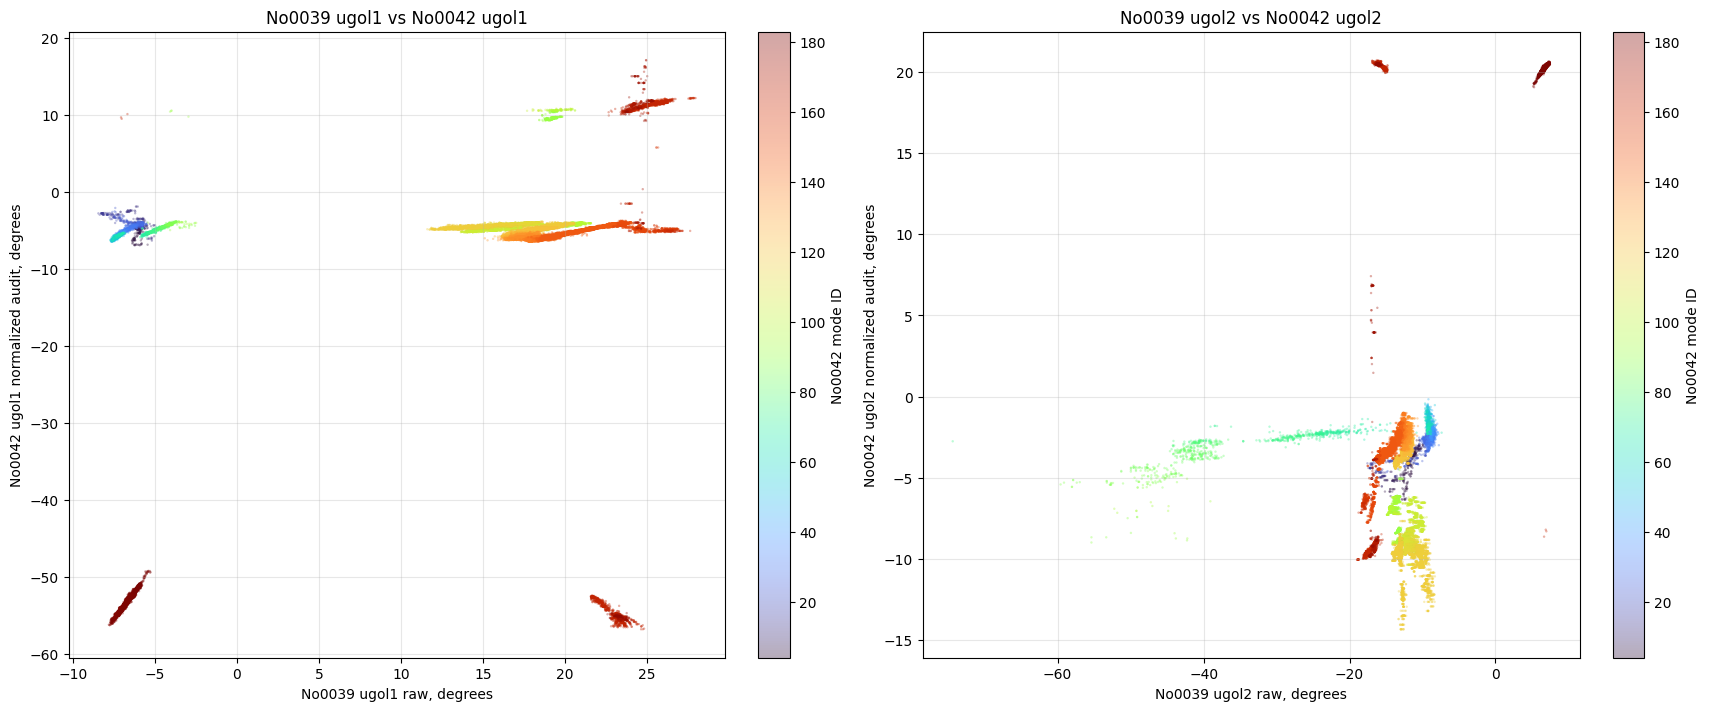

ANGLE CORRELATION SUMMARY


,comparison,pearson_r,n_pairs
0,ugol1: No0039 raw vs No0042 audit,0.670462,50709
1,ugol2: No0039 raw vs No0042 audit,0.728314,50709


In [ ]:
df_scatter = (
    df_angle_compare
    .loc[
        df_angle_compare[
            "angle0042NormalizedAvailable"
        ]
        .fillna(False)
        .astype(bool)
    ]
    .copy()
)

figure, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(17, 7),
    constrained_layout=True,
)


scatter_ugol1 = axes[0].scatter(
    df_scatter["ugol1DegRaw0039"],
    df_scatter["ugol1DegNorm0042"],
    c=df_scatter["angle0042ModeId"],
    cmap="turbo",
    s=3,
    alpha=0.35,
    linewidths=0.0,
)

axes[0].set_title(
    "No0039 ugol1 vs No0042 ugol1"
)

axes[0].set_xlabel(
    "No0039 ugol1 raw, degrees"
)

axes[0].set_ylabel(
    "No0042 ugol1 normalized audit, degrees"
)

axes[0].grid(
    True,
    alpha=0.30,
)

figure.colorbar(
    scatter_ugol1,
    ax=axes[0],
    label="No0042 mode ID",
)


scatter_ugol2 = axes[1].scatter(
    df_scatter["ugol2DegRaw0039"],
    df_scatter["ugol2DegNorm0042"],
    c=df_scatter["angle0042ModeId"],
    cmap="turbo",
    s=3,
    alpha=0.35,
    linewidths=0.0,
)

axes[1].set_title(
    "No0039 ugol2 vs No0042 ugol2"
)

axes[1].set_xlabel(
    "No0039 ugol2 raw, degrees"
)

axes[1].set_ylabel(
    "No0042 ugol2 normalized audit, degrees"
)

axes[1].grid(
    True,
    alpha=0.30,
)

figure.colorbar(
    scatter_ugol2,
    ax=axes[1],
    label="No0042 mode ID",
)

plt.show()


correlation_table = pd.DataFrame(
    {
        "comparison": [
            "ugol1: No0039 raw vs No0042 audit",
            "ugol2: No0039 raw vs No0042 audit",
        ],
        "pearson_r": [
            df_scatter[
                [
                    "ugol1DegRaw0039",
                    "ugol1DegNorm0042",
                ]
            ]
            .corr()
            .iloc[0, 1],
            df_scatter[
                [
                    "ugol2DegRaw0039",
                    "ugol2DegNorm0042",
                ]
            ]
            .corr()
            .iloc[0, 1],
        ],
        "n_pairs": [
            int(
                df_scatter[
                    [
                        "ugol1DegRaw0039",
                        "ugol1DegNorm0042",
                    ]
                ]
                .dropna()
                .shape[0]
            ),
            int(
                df_scatter[
                    [
                        "ugol2DegRaw0039",
                        "ugol2DegNorm0042",
                    ]
                ]
                .dropna()
                .shape[0]
            ),
        ],
    }
)

print("ANGLE CORRELATION SUMMARY")
display(correlation_table)

In [ ]:
%%writefile -a /content/hoarfrost_project/src/angle_normalization.py


# ---------------------------------------------------------------------------
# Automatic methodology extension.
#
# This extension implements the original requested methodology:
# mode segmentation -> reference mode -> best transform selection
# -> offset / sign flips / axis swap -> normalized ugol1 / ugol2.
# ---------------------------------------------------------------------------

_original_validate_angle_normalization_config = (
    _validate_config
)

_original_normalize_sensor_angles = (
    normalize_sensor_angles
)


def _validate_config(
    config: AngleNormalizationConfig,
) -> None:
    allowed_modes = {
        "disabled",
        "audit_only",
        "approved_offsets_only",
        "automatic_methodology",
    }

    if config.mode not in allowed_modes:
        raise ValueError(
            "Unsupported angle normalization mode: "
            f"{config.mode!r}. "
            f"Allowed modes: {sorted(allowed_modes)}"
        )

    if config.max_continuity_gap_seconds <= 0.0:
        raise ValueError(
            "max_continuity_gap_seconds must be positive."
        )

    if config.sustained_shift_threshold_deg <= 0.0:
        raise ValueError(
            "sustained_shift_threshold_deg must be positive."
        )

    if config.min_sustained_points < 2:
        raise ValueError(
            "min_sustained_points must be at least 2."
        )

    if config.local_window_points < 1:
        raise ValueError(
            "local_window_points must be at least 1."
        )

    if config.reference_mode_strategy not in {
        "first",
        "largest",
    }:
        raise ValueError(
            "reference_mode_strategy must be "
            "'first' or 'largest'."
        )


def _estimate_automatic_methodology_transforms(
    dataframe: pd.DataFrame,
    modes: pd.DataFrame,
) -> pd.DataFrame:
    if dataframe.empty or modes.empty:
        return pd.DataFrame(
            columns=[
                "angle_mode_id",
                "reference_mode_id",
                "transform",
                "sign_ugol1",
                "sign_ugol2",
                "swap_axes",
                "offset_ugol1_deg",
                "offset_ugol2_deg",
                "residual_jump_deg",
                "confidence",
                "transform_status",
            ]
        )

    reference_mode_id = int(
        modes["reference_mode_id"].iloc[0]
    )

    reference_rows = dataframe.loc[
        dataframe["angle_mode_id"].eq(
            reference_mode_id
        )
        & dataframe["angles_available"]
    ].copy()

    if reference_rows.empty:
        raise RuntimeError(
            "Automatic angle normalization cannot "
            "estimate the reference mode because "
            "the reference mode has no valid "
            "ugol1/ugol2 pairs."
        )

    reference_median = np.array(
        [
            float(
                reference_rows[
                    "ugol1_raw_deg"
                ].median()
            ),
            float(
                reference_rows[
                    "ugol2_raw_deg"
                ].median()
            ),
        ]
    )

    transform_candidates = [
        {
            "transform": "offset",
            "sign_ugol1": 1,
            "sign_ugol2": 1,
            "swap_axes": False,
        },
        {
            "transform": "sign_flip_ugol1",
            "sign_ugol1": -1,
            "sign_ugol2": 1,
            "swap_axes": False,
        },
        {
            "transform": "sign_flip_ugol2",
            "sign_ugol1": 1,
            "sign_ugol2": -1,
            "swap_axes": False,
        },
        {
            "transform": "sign_flip_both",
            "sign_ugol1": -1,
            "sign_ugol2": -1,
            "swap_axes": False,
        },
        {
            "transform": "swap_axes",
            "sign_ugol1": 1,
            "sign_ugol2": 1,
            "swap_axes": True,
        },
    ]

    records = []

    for _, mode in modes.iterrows():
        mode_id = int(mode["angle_mode_id"])

        mode_rows = dataframe.loc[
            dataframe["angle_mode_id"].eq(
                mode_id
            )
            & dataframe["angles_available"]
        ].copy()

        if mode_rows.empty:
            continue

        mode_median = np.array(
            [
                float(
                    mode_rows[
                        "ugol1_raw_deg"
                    ].median()
                ),
                float(
                    mode_rows[
                        "ugol2_raw_deg"
                    ].median()
                ),
            ]
        )

        best_record = None

        for candidate in transform_candidates:
            if candidate["swap_axes"]:
                transformed_median = np.array(
                    [
                        mode_median[1],
                        mode_median[0],
                    ]
                )
            else:
                transformed_median = np.array(
                    [
                        candidate["sign_ugol1"],
                        candidate["sign_ugol2"],
                    ],
                    dtype=float,
                ) * mode_median

            residual_jump = float(
                np.linalg.norm(
                    transformed_median
                    - reference_median
                )
            )

            if (
                best_record is None
                or residual_jump
                < best_record["residual_jump_deg"]
            ):
                offset_vector = (
                    transformed_median
                    - reference_median
                )

                if residual_jump < 2.0:
                    confidence = 0.95
                elif residual_jump < 5.0:
                    confidence = 0.80
                elif residual_jump < 10.0:
                    confidence = 0.60
                else:
                    confidence = 0.40

                best_record = {
                    "angle_mode_id": mode_id,
                    "reference_mode_id": (
                        reference_mode_id
                    ),
                    "transform": (
                        candidate["transform"]
                    ),
                    "sign_ugol1": int(
                        candidate["sign_ugol1"]
                    ),
                    "sign_ugol2": int(
                        candidate["sign_ugol2"]
                    ),
                    "swap_axes": bool(
                        candidate["swap_axes"]
                    ),
                    "offset_ugol1_deg": float(
                        offset_vector[0]
                    ),
                    "offset_ugol2_deg": float(
                        offset_vector[1]
                    ),
                    "residual_jump_deg": (
                        residual_jump
                    ),
                    "confidence": float(
                        confidence
                    ),
                    "transform_status": (
                        "automatic_methodology_applied"
                    ),
                }

        records.append(best_record)

    return pd.DataFrame(records)


def _apply_automatic_methodology_transforms(
    dataframe: pd.DataFrame,
    transforms: pd.DataFrame,
) -> pd.DataFrame:
    result = dataframe.copy()

    result["ugol1_norm_deg"] = result[
        "ugol1_raw_deg"
    ]

    result["ugol2_norm_deg"] = result[
        "ugol2_raw_deg"
    ]

    result["angle_transform"] = "identity"
    result["angle_offset_ugol1_deg"] = 0.0
    result["angle_offset_ugol2_deg"] = 0.0
    result["angle_normalization_approved"] = False
    result["angle_normalization_automatic"] = False
    result["angle_normalization_quality"] = (
        "automatic_methodology_unassigned"
    )

    if transforms.empty:
        result["angle_normalization_quality"] = (
            "automatic_methodology_no_transform"
        )
        return result

    for _, transform in transforms.iterrows():
        mode_id = int(
            transform["angle_mode_id"]
        )

        mask = result["angle_mode_id"].eq(
            mode_id
        )

        raw_ugol1 = pd.to_numeric(
            result.loc[
                mask,
                "ugol1_raw_deg",
            ],
            errors="coerce",
        )

        raw_ugol2 = pd.to_numeric(
            result.loc[
                mask,
                "ugol2_raw_deg",
            ],
            errors="coerce",
        )

        if bool(transform["swap_axes"]):
            ugol1_temp = raw_ugol2
            ugol2_temp = raw_ugol1
        else:
            ugol1_temp = raw_ugol1
            ugol2_temp = raw_ugol2

        result.loc[
            mask,
            "ugol1_norm_deg",
        ] = (
            float(transform["sign_ugol1"])
            * ugol1_temp
            - float(
                transform[
                    "offset_ugol1_deg"
                ]
            )
        )

        result.loc[
            mask,
            "ugol2_norm_deg",
        ] = (
            float(transform["sign_ugol2"])
            * ugol2_temp
            - float(
                transform[
                    "offset_ugol2_deg"
                ]
            )
        )

        result.loc[
            mask,
            "angle_transform",
        ] = str(
            transform["transform"]
        )

        result.loc[
            mask,
            "angle_offset_ugol1_deg",
        ] = float(
            transform["offset_ugol1_deg"]
        )

        result.loc[
            mask,
            "angle_offset_ugol2_deg",
        ] = float(
            transform["offset_ugol2_deg"]
        )

        result.loc[
            mask,
            "angle_normalization_automatic",
        ] = True

        result.loc[
            mask,
            "angle_normalization_quality",
        ] = (
            "automatic_methodology_applied"
        )

    return result


def normalize_sensor_angles(
    dataframe: pd.DataFrame,
    config: AngleNormalizationConfig = (
        AngleNormalizationConfig()
    ),
    timestamp_column: str = "created_at",
    ugol1_column: str = "ugol1",
    ugol2_column: str = "ugol2",
) -> Dict[str, Any]:
    if config.mode != "automatic_methodology":
        return _original_normalize_sensor_angles(
            dataframe=dataframe,
            config=config,
            timestamp_column=timestamp_column,
            ugol1_column=ugol1_column,
            ugol2_column=ugol2_column,
        )

    _validate_config(config)

    audit_config = AngleNormalizationConfig(
        sensor_id=config.sensor_id,
        max_continuity_gap_seconds=(
            config.max_continuity_gap_seconds
        ),
        sustained_shift_threshold_deg=(
            config.sustained_shift_threshold_deg
        ),
        min_sustained_points=(
            config.min_sustained_points
        ),
        local_window_points=(
            config.local_window_points
        ),
        transition_merge_seconds=(
            config.transition_merge_seconds
        ),
        min_mode_points=config.min_mode_points,
        min_mode_duration_seconds=(
            config.min_mode_duration_seconds
        ),
        reference_mode_strategy=(
            config.reference_mode_strategy
        ),
        mode="audit_only",
        approved_offsets={},
    )

    result = _original_normalize_sensor_angles(
        dataframe=dataframe,
        config=audit_config,
        timestamp_column=timestamp_column,
        ugol1_column=ugol1_column,
        ugol2_column=ugol2_column,
    )

    transforms = (
        _estimate_automatic_methodology_transforms(
            dataframe=result["normalized"],
            modes=result["modes"],
        )
    )

    normalized = (
        _apply_automatic_methodology_transforms(
            dataframe=result["normalized"],
            transforms=transforms,
        )
    )

    summary = dict(result["summary"])

    summary.update(
        {
            "mode": "automatic_methodology",
            "n_automatic_transform_modes": int(
                len(transforms)
            ),
            "n_automatic_transform_rows": int(
                normalized[
                    "angle_normalization_automatic"
                ]
                .sum()
            ),
            "n_automatic_offset_rows": int(
                normalized[
                    "angle_transform"
                ]
                .eq("offset")
                .sum()
            ),
            "n_automatic_sign_flip_ugol1_rows": int(
                normalized[
                    "angle_transform"
                ]
                .eq("sign_flip_ugol1")
                .sum()
            ),
            "n_automatic_sign_flip_ugol2_rows": int(
                normalized[
                    "angle_transform"
                ]
                .eq("sign_flip_ugol2")
                .sum()
            ),
            "n_automatic_sign_flip_both_rows": int(
                normalized[
                    "angle_transform"
                ]
                .eq("sign_flip_both")
                .sum()
            ),
            "n_automatic_swap_axes_rows": int(
                normalized[
                    "angle_transform"
                ]
                .eq("swap_axes")
                .sum()
            ),
        }
    )

    return {
        "normalized": normalized,
        "shift_candidates": result[
            "shift_candidates"
        ],
        "modes": result["modes"],
        "offset_candidates": transforms,
        "summary": summary,
    }

Appending to /content/hoarfrost_project/src/angle_normalization.py


In [ ]:
%%writefile -a /content/hoarfrost_project/src/data_normalization.py


# ---------------------------------------------------------------------------
# Full strict No0042 replacement extension.
#
# automatic_methodology:
#   normalized No0042 ugol1/ugol2 become the only active angle source.
#   Legacy No0039 is preserved only in explicit *_0039 provenance columns.
# ---------------------------------------------------------------------------

_original_validate_angle0042_integration_config = (
    _validate_angle0042_integration_config
)

_original_attach_optional_normalized_angles_0042 = (
    attach_optional_normalized_angles_0042
)


def _validate_angle0042_integration_config(
    config: Angle0042IntegrationConfig,
) -> None:
    allowed_modes = {
        "disabled",
        "audit_only",
        "approved_offsets_only",
        "automatic_methodology",
    }

    if config.max_angle_age_seconds <= 0.0:
        raise ValueError(
            "max_angle_age_seconds must be positive."
        )

    if config.normalization_mode not in allowed_modes:
        raise ValueError(
            "Unsupported No0042 normalization mode: "
            f"{config.normalization_mode!r}."
        )

    if (
        config.use_normalized_0042_as_active_angles
        and not config.enabled
    ):
        raise ValueError(
            "No0042 active-angle substitution requires "
            "enabled=True."
        )

    allowed_active_modes = {
        "approved_offsets_only",
        "automatic_methodology",
    }

    if (
        config.use_normalized_0042_as_active_angles
        and config.normalization_mode
        not in allowed_active_modes
    ):
        raise ValueError(
            "Active No0042 substitution requires "
            "normalization_mode to be either "
            "'approved_offsets_only' or "
            "'automatic_methodology'."
        )


def attach_optional_normalized_angles_0042(
    normalized_dataframe: pd.DataFrame,
    sensor_angle_0042_csv_path: str | Path,
    config: Angle0042IntegrationConfig,
) -> NormalizationResult:
    result = (
        _original_attach_optional_normalized_angles_0042(
            normalized_dataframe=normalized_dataframe,
            sensor_angle_0042_csv_path=(
                sensor_angle_0042_csv_path
            ),
            config=config,
        )
    )

    if not (
        config.enabled
        and config.use_normalized_0042_as_active_angles
        and config.normalization_mode
        == "automatic_methodology"
    ):
        return result

    dataframe = result.dataframe.copy()

    required_columns = [
        "ugol1DegNorm0042",
        "ugol2DegNorm0042",
        "angle0042NormalizedAvailable",
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in dataframe.columns
    ]

    if missing_columns:
        raise KeyError(
            "Automatic No0042 replacement requires "
            "columns: "
            f"{missing_columns}"
        )

    active_valid = (
        dataframe[
            "angle0042NormalizedAvailable"
        ]
        .fillna(False)
        .astype(bool)
    )

    dataframe["ugol1DegRaw"] = pd.to_numeric(
        dataframe["ugol1DegNorm0042"],
        errors="coerce",
    ).where(active_valid)

    dataframe["ugol2DegRaw"] = pd.to_numeric(
        dataframe["ugol2DegNorm0042"],
        errors="coerce",
    ).where(active_valid)

    dataframe["rawAnglesAvailable"] = active_valid

    dataframe["rawAngleSource"] = np.where(
        active_valid,
        (
            "Sensor-VL-module-3-No0042:"
            "automatic_methodology_normalized"
        ),
        (
            "Sensor-VL-module-3-No0042:"
            "unavailable_or_stale"
        ),
    )

    dataframe["rawAngleFieldsVersion"] = (
        "angle0042_automatic_methodology_active_v1"
    )

    dataframe["angle0042UsedAsActiveSource"] = True

    dataframe["activeAngleSourcePolicy"] = (
        "normalized_no0042_strict"
    )

    dataframe["angle0042AutomaticMethodologyApplied"] = (
        active_valid
    )

    provenance = dict(result.provenance)

    provenance.update(
        {
            "angle0042_used_as_active_source": True,
            "active_angle_source_policy": (
                "normalized_no0042_strict"
            ),
            "angle0042_automatic_methodology": True,
            "n_angle0042_automatic_active_rows": int(
                active_valid.sum()
            ),
            "n_angle0042_active_unavailable_rows": int(
                (~active_valid).sum()
            ),
        }
    )

    dataframe.attrs.update(provenance)

    return NormalizationResult(
        dataframe=dataframe,
        provenance=provenance,
    )

Appending to /content/hoarfrost_project/src/data_normalization.py


In [ ]:
import importlib
import sys


for module_name in list(sys.modules):
    if (
        module_name == "src"
        or module_name.startswith("src.")
    ):
        del sys.modules[module_name]

importlib.invalidate_caches()


from src.angle_normalization import (
    AngleNormalizationConfig,
    normalize_sensor_angles,
)

from src.data_normalization import (
    Angle0042IntegrationConfig,
    build_canonical_dataset_with_optional_angle_0042,
)


print(
    "Automatic No0042 methodology import passed."
)

print(
    "Angle module:",
    normalize_sensor_angles,
)

print(
    "No0042 canonical builder:",
    build_canonical_dataset_with_optional_angle_0042,
)

Automatic No0042 methodology import passed.
Angle module: <function normalize_sensor_angles at 0x7b167ff51300>
No0042 canonical builder: <function build_canonical_dataset_with_optional_angle_0042 at 0x7b167ff36fc0>


In [ ]:
import numpy as np
import pandas as pd


required_strict_columns = [
    "ugol1DegRaw",
    "ugol2DegRaw",
    "ugol1DegRaw0039",
    "ugol2DegRaw0039",
    "ugol1DegNorm0042",
    "ugol2DegNorm0042",
    "angle0042RawAvailable",
    "angle0042NormalizedAvailable",
    "angle0042UsedAsActiveSource",
    "angle0042NormalizationQuality",
    "rawAnglesAvailable",
    "rawAngleSource",
    "activeAngleSourcePolicy",
]

missing_strict_columns = [
    column
    for column in required_strict_columns
    if column not in df_norm.columns
]

assert not missing_strict_columns, (
    "Strict No0042 integration fields are missing: "
    f"{missing_strict_columns}"
)


assert (
    normalization_provenance[
        "angle0042_enabled"
    ]
    is True
)

assert (
    normalization_provenance[
        "angle0042_normalization_mode"
    ]
    == "automatic_methodology"
)

assert (
    normalization_provenance[
        "angle0042_used_as_active_source"
    ]
    is True
)

assert (
    normalization_provenance[
        "active_angle_source_policy"
    ]
    == "normalized_no0042_strict"
)


active_mask = (
    df_norm[
        "rawAnglesAvailable"
    ]
    .fillna(False)
    .astype(bool)
)

no0042_valid_mask = (
    df_norm[
        "angle0042NormalizedAvailable"
    ]
    .fillna(False)
    .astype(bool)
)

assert active_mask.equals(
    no0042_valid_mask
), (
    "Active rawAnglesAvailable must exactly match "
    "No0042 normalized availability in strict mode."
)


ugol1_active_equals_no0042 = np.allclose(
    pd.to_numeric(
        df_norm.loc[
            active_mask,
            "ugol1DegRaw",
        ],
        errors="coerce",
    ),
    pd.to_numeric(
        df_norm.loc[
            active_mask,
            "ugol1DegNorm0042",
        ],
        errors="coerce",
    ),
    equal_nan=True,
)

ugol2_active_equals_no0042 = np.allclose(
    pd.to_numeric(
        df_norm.loc[
            active_mask,
            "ugol2DegRaw",
        ],
        errors="coerce",
    ),
    pd.to_numeric(
        df_norm.loc[
            active_mask,
            "ugol2DegNorm0042",
        ],
        errors="coerce",
    ),
    equal_nan=True,
)

assert ugol1_active_equals_no0042
assert ugol2_active_equals_no0042


active_sources = (
    df_norm[
        "rawAngleSource"
    ]
    .astype("string")
)

no0039_fallback_rows = int(
    active_mask
    & active_sources.str.contains(
        "No0039",
        na=False,
    )
).sum()

assert no0039_fallback_rows == 0, (
    "Strict No0042 mode must not use No0039 "
    "as an active fallback source."
)


print("STRICT NO0042 ACTIVE-ANGLE VALIDATION")
print("=" * 78)

print(
    "Policy:",
    normalization_provenance[
        "active_angle_source_policy"
    ],
)

print(
    "Active No0042 angle rows:",
    int(active_mask.sum()),
)

print(
    "No0042 unavailable angle rows:",
    int((~active_mask).sum()),
)

print(
    "Active ugol1 equals normalized No0042:",
    ugol1_active_equals_no0042,
)

print(
    "Active ugol2 equals normalized No0042:",
    ugol2_active_equals_no0042,
)

print(
    "No0039 active fallback rows:",
    no0039_fallback_rows,
)

print(
    "\nActive raw-angle source counts:"
)

display(
    df_norm[
        "rawAngleSource"
    ]
    .astype("string")
    .value_counts(
        dropna=False,
    )
    .rename("count")
    .to_frame()
)


print(
    "\nNo0042 transform distribution:"
)

display(
    df_norm[
        "angle0042Transform"
    ]
    .astype("string")
    .value_counts(
        dropna=False,
    )
    .rename("count")
    .to_frame()
)


print(
    "\nNo0042 normalization-quality distribution:"
)

display(
    df_norm[
        "angle0042NormalizationQuality"
    ]
    .astype("string")
    .value_counts(
        dropna=False,
    )
    .rename("count")
    .to_frame()
)

TypeError: cannot convert the series to <class 'int'>

In [ ]:
from pathlib import Path


STRICT_OUTPUT_DIR = (
    PROJECT_ROOT
    / "output_angle0042_auto_strict"
)

STRICT_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


required_runtime_objects = [
    "df_norm",
    "df_cal",
    "df_sim",
    "df_provenance",
    "df_goryachev_reference_raw",
    "df_goryachev_reference_clean",
    "df_goryachev_reference_states",
    "mechanical_events",
    "mechanical_event_meteo_audit",
    "input_quality_rows",
    "input_quality_intervals",
    "model_quality_intervals",
    "mechanical_event_input_quality",
    "input_quality_summary_table",
    "reference_quality_summary",
    "reference_candidate_rows",
    "reference_quality_rows",
    "strict_physics_set",
    "review_sensitivity_set",
    "reference_unverified_set",
]

missing_runtime_objects = [
    object_name
    for object_name in required_runtime_objects
    if object_name not in globals()
]

assert not missing_runtime_objects, (
    "Cannot snapshot strict experiment. "
    "Missing objects: "
    f"{missing_runtime_objects}"
)


strict_output_files = {
    "normalized_dataset_canonical.csv": df_norm,
    "calibrated_dataset_full.csv": df_cal,
    "simulation_results_full.csv": df_sim,
    "pipeline_provenance.csv": df_provenance,
    "goryachev_no_ice_reference_raw.csv": (
        df_goryachev_reference_raw
    ),
    "goryachev_no_ice_reference_clean.csv": (
        df_goryachev_reference_clean
    ),
    "goryachev_fixed_reference_states.csv": (
        df_goryachev_reference_states
    ),
    "mechanical_events.csv": mechanical_events,
    "mechanical_event_meteo_audit.csv": (
        mechanical_event_meteo_audit
    ),
    "input_quality_rows.csv": input_quality_rows,
    "input_quality_intervals.csv": (
        input_quality_intervals
    ),
    "model_quality_intervals.csv": (
        model_quality_intervals
    ),
    "mechanical_event_input_quality.csv": (
        mechanical_event_input_quality
    ),
    "input_quality_summary.csv": (
        input_quality_summary_table
    ),
    "goryachev_reference_label_quality.csv": (
        reference_quality_summary
    ),
    "goryachev_reference_candidate_rows.csv": (
        reference_candidate_rows
    ),
    "mechanical_reference_quality_rows.csv": (
        reference_quality_rows
    ),
    "makkonen_goryachev_strict_physics_set.csv": (
        strict_physics_set
    ),
    "makkonen_goryachev_review_sensitivity_set.csv": (
        review_sensitivity_set
    ),
    "makkonen_goryachev_reference_unverified_set.csv": (
        reference_unverified_set
    ),
}


for filename, dataframe in strict_output_files.items():
    output_path = STRICT_OUTPUT_DIR / filename

    dataframe.to_csv(
        output_path,
        index=False,
    )

    assert output_path.exists(), (
        f"Strict artifact was not saved: "
        f"{output_path}"
    )

    assert output_path.stat().st_size > 0, (
        f"Strict artifact is empty: "
        f"{output_path}"
    )


print("STRICT NO0042 EXPERIMENT SNAPSHOT SAVED")
print("=" * 78)

print(
    "Directory:",
    STRICT_OUTPUT_DIR,
)

for filename in strict_output_files:
    print(
        STRICT_OUTPUT_DIR / filename
    )

STRICT NO0042 EXPERIMENT SNAPSHOT SAVED
Directory: /content/hoarfrost_project/output_angle0042_auto_strict
/content/hoarfrost_project/output_angle0042_auto_strict/normalized_dataset_canonical.csv
/content/hoarfrost_project/output_angle0042_auto_strict/calibrated_dataset_full.csv
/content/hoarfrost_project/output_angle0042_auto_strict/simulation_results_full.csv
/content/hoarfrost_project/output_angle0042_auto_strict/pipeline_provenance.csv
/content/hoarfrost_project/output_angle0042_auto_strict/goryachev_no_ice_reference_raw.csv
/content/hoarfrost_project/output_angle0042_auto_strict/goryachev_no_ice_reference_clean.csv
/content/hoarfrost_project/output_angle0042_auto_strict/goryachev_fixed_reference_states.csv
/content/hoarfrost_project/output_angle0042_auto_strict/mechanical_events.csv
/content/hoarfrost_project/output_angle0042_auto_strict/mechanical_event_meteo_audit.csv
/content/hoarfrost_project/output_angle0042_auto_strict/input_quality_rows.csv
/content/hoarfrost_project/output

In [ ]:
import numpy as np
import pandas as pd


active_mask = (
    df_norm[
        "rawAnglesAvailable"
    ]
    .fillna(False)
    .astype(bool)
)

no0042_valid_mask = (
    df_norm[
        "angle0042NormalizedAvailable"
    ]
    .fillna(False)
    .astype(bool)
)

active_sources = (
    df_norm[
        "rawAngleSource"
    ]
    .astype("string")
)


assert (
    normalization_provenance[
        "active_angle_source_policy"
    ]
    == "normalized_no0042_strict"
)

assert active_mask.equals(
    no0042_valid_mask
)


ugol1_active_equals_no0042 = np.allclose(
    pd.to_numeric(
        df_norm.loc[
            active_mask,
            "ugol1DegRaw",
        ],
        errors="coerce",
    ),
    pd.to_numeric(
        df_norm.loc[
            active_mask,
            "ugol1DegNorm0042",
        ],
        errors="coerce",
    ),
    equal_nan=True,
)

ugol2_active_equals_no0042 = np.allclose(
    pd.to_numeric(
        df_norm.loc[
            active_mask,
            "ugol2DegRaw",
        ],
        errors="coerce",
    ),
    pd.to_numeric(
        df_norm.loc[
            active_mask,
            "ugol2DegNorm0042",
        ],
        errors="coerce",
    ),
    equal_nan=True,
)

assert ugol1_active_equals_no0042
assert ugol2_active_equals_no0042


no0039_fallback_rows = int(
    (
        active_mask
        & active_sources.str.contains(
            "No0039",
            na=False,
        )
    )
    .sum()
)

assert no0039_fallback_rows == 0


print("STRICT NO0042 ACTIVE-ANGLE VALIDATION")
print("=" * 78)

print(
    "Policy:",
    normalization_provenance[
        "active_angle_source_policy"
    ],
)

print(
    "Active No0042 rows:",
    int(active_mask.sum()),
)

print(
    "Unavailable active-angle rows:",
    int((~active_mask).sum()),
)

print(
    "ugol1 active == No0042 normalized:",
    ugol1_active_equals_no0042,
)

print(
    "ugol2 active == No0042 normalized:",
    ugol2_active_equals_no0042,
)

print(
    "No0039 active fallback rows:",
    no0039_fallback_rows,
)

print("\nActive angle-source counts:")

display(
    active_sources
    .value_counts(
        dropna=False,
    )
    .rename("count")
    .to_frame()
)

print("\nNo0042 transform distribution:")

display(
    df_norm[
        "angle0042Transform"
    ]
    .astype("string")
    .value_counts(
        dropna=False,
    )
    .rename("count")
    .to_frame()
)

STRICT NO0042 ACTIVE-ANGLE VALIDATION
Policy: normalized_no0042_strict
Active No0042 rows: 50709
Unavailable active-angle rows: 5685
ugol1 active == No0042 normalized: True
ugol2 active == No0042 normalized: True
No0039 active fallback rows: 0

Active angle-source counts:


,count
rawAngleSource,
Sensor-VL-module-3-No0042:automatic_methodology_normalized,50709
Sensor-VL-module-3-No0042:unavailable_or_stale,5685



No0042 transform distribution:


,count
angle0042Transform,
offset,38284
swap_axes,9927
sign_flip_ugol2,6320
sign_flip_ugol1,1846
sign_flip_both,15
<NA>,2


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


# ---------------------------------------------------------------------
# 1. Validate required columns.
# ---------------------------------------------------------------------

required_norm_columns = [
    "timestamp",
    "ugol1DegRaw",
    "ugol2DegRaw",
    "ugol1DegNorm0042",
    "ugol2DegNorm0042",
    "angle0042Transform",
    "angle0042ModeId",
    "angle0042NormalizedAvailable",
    "rawAnglesAvailable",
    "rawAngleSource",
    "activeAngleSourcePolicy",
]

required_cal_columns = [
    "timestamp",
    "phiHdeg",
    "phiK1deg",
    "isNoIceReference",
]

required_sim_columns = [
    "timestamp",
    "gorCm",
    "gorStatus",
]

missing_norm_columns = [
    column
    for column in required_norm_columns
    if column not in df_norm.columns
]

missing_cal_columns = [
    column
    for column in required_cal_columns
    if column not in df_cal.columns
]

missing_sim_columns = [
    column
    for column in required_sim_columns
    if column not in df_sim.columns
]

assert not missing_norm_columns, (
    "df_norm is missing columns: "
    f"{missing_norm_columns}"
)

assert not missing_cal_columns, (
    "df_cal is missing columns: "
    f"{missing_cal_columns}"
)

assert not missing_sim_columns, (
    "df_sim is missing columns: "
    f"{missing_sim_columns}"
)


# ---------------------------------------------------------------------
# 2. Build strict No0042 analysis table.
# ---------------------------------------------------------------------

norm_columns = [
    column
    for column in [
        "timestamp",
        "ugol1DegRaw",
        "ugol2DegRaw",
        "ugol1DegRaw0039",
        "ugol2DegRaw0039",
        "ugol1DegNorm0042",
        "ugol2DegNorm0042",
        "angle0042Transform",
        "angle0042ModeId",
        "angle0042NormalizedAvailable",
        "rawAnglesAvailable",
        "rawAngleSource",
        "activeAngleSourcePolicy",
    ]
    if column in df_norm.columns
]

cal_columns = [
    "timestamp",
    "phiHdeg",
    "phiK1deg",
    "isNoIceReference",
]

sim_columns = [
    column
    for column in [
        "timestamp",
        "gorCm",
        "gorStatus",
        "gorFgN",
        "gorDeltaFgN",
        "gorSagM",
        "mechanicalEventId",
    ]
    if column in df_sim.columns
]


df_norm_plot = (
    df_norm[norm_columns]
    .copy()
)

df_cal_plot = (
    df_cal[cal_columns]
    .copy()
)

df_sim_plot = (
    df_sim[sim_columns]
    .copy()
)


for dataframe in [
    df_norm_plot,
    df_cal_plot,
    df_sim_plot,
]:
    dataframe["timestamp"] = pd.to_datetime(
        dataframe["timestamp"],
        errors="coerce",
    )

    dataframe.dropna(
        subset=["timestamp"],
        inplace=True,
    )

    dataframe.sort_values(
        "timestamp",
        inplace=True,
    )

    dataframe.drop_duplicates(
        subset=["timestamp"],
        keep="last",
        inplace=True,
    )


assert df_norm_plot["timestamp"].is_unique
assert df_cal_plot["timestamp"].is_unique
assert df_sim_plot["timestamp"].is_unique


df_strict_plot = (
    df_norm_plot
    .merge(
        df_cal_plot,
        on="timestamp",
        how="left",
        validate="one_to_one",
    )
    .merge(
        df_sim_plot,
        on="timestamp",
        how="left",
        validate="one_to_one",
    )
    .sort_values("timestamp")
    .reset_index(drop=True)
)


numeric_columns = [
    "ugol1DegRaw",
    "ugol2DegRaw",
    "ugol1DegNorm0042",
    "ugol2DegNorm0042",
    "ugol1DegRaw0039",
    "ugol2DegRaw0039",
    "phiHdeg",
    "phiK1deg",
    "gorCm",
    "gorFgN",
    "gorDeltaFgN",
    "gorSagM",
]

for column in numeric_columns:
    if column in df_strict_plot.columns:
        df_strict_plot[column] = pd.to_numeric(
            df_strict_plot[column],
            errors="coerce",
        )


df_strict_plot["gorCmMm"] = (
    df_strict_plot["gorCm"]
    * 1000.0
)

df_strict_plot["activeAnglesAvailable"] = (
    df_strict_plot["rawAnglesAvailable"]
    .fillna(False)
    .astype(bool)
)

df_strict_plot["isNoIceReference"] = (
    df_strict_plot["isNoIceReference"]
    .fillna(False)
    .astype(bool)
)

df_strict_plot["gorStatus"] = (
    df_strict_plot["gorStatus"]
    .astype("string")
)


gor_ok_mask = (
    df_strict_plot["gorStatus"]
    .eq("ok")
    & df_strict_plot["gorCmMm"].notna()
)

gor_no_ice_mask = (
    df_strict_plot["gorStatus"]
    .eq("no_ice")
)

gor_out_of_range_mask = (
    df_strict_plot["gorStatus"]
    .eq("angle_out_of_range")
)

gor_no_reference_mask = (
    df_strict_plot["gorStatus"]
    .eq("no_reference_for_raw_angle_segment")
)

no0042_unavailable_mask = (
    ~df_strict_plot[
        "activeAnglesAvailable"
    ]
)

no_ice_reference_mask = (
    df_strict_plot[
        "isNoIceReference"
    ]
)


# ---------------------------------------------------------------------
# 3. Diagnostic summary.
# ---------------------------------------------------------------------

print("STRICT NO0042 GORYACHEV DIAGNOSTIC SUMMARY")
print("=" * 78)

print(
    "Active angle source policy:",
    df_strict_plot[
        "activeAngleSourcePolicy"
    ]
    .dropna()
    .unique()
    .tolist(),
)

print(
    "Rows:",
    len(df_strict_plot),
)

print(
    "Rows with active No0042 angles:",
    int(
        df_strict_plot[
            "activeAnglesAvailable"
        ].sum()
    ),
)

print(
    "Rows without active No0042 angles:",
    int(
        no0042_unavailable_mask.sum()
    ),
)

print(
    "Goryachev ok rows:",
    int(gor_ok_mask.sum()),
)

print(
    "Goryachev angle_out_of_range rows:",
    int(gor_out_of_range_mask.sum()),
)

print(
    "Goryachev no-reference rows:",
    int(gor_no_reference_mask.sum()),
)

print(
    "No-ice reference rows:",
    int(no_ice_reference_mask.sum()),
)

print(
    "Maximum Goryachev c_m, mm:",
    round(
        float(
            df_strict_plot.loc[
                gor_ok_mask,
                "gorCmMm",
            ].max()
        ),
        3,
    ),
)


max_cm_row = (
    df_strict_plot
    .loc[gor_ok_mask]
    .sort_values(
        "gorCmMm",
        ascending=False,
    )
    .head(1)
    .copy()
)

print("\nMAXIMUM GORYACHEV THICKNESS ROW")
display(
    max_cm_row[
        [
            column
            for column in [
                "timestamp",
                "gorCmMm",
                "gorStatus",
                "gorFgN",
                "gorDeltaFgN",
                "gorSagM",
                "phiHdeg",
                "phiK1deg",
                "ugol1DegRaw",
                "ugol2DegRaw",
                "ugol1DegNorm0042",
                "ugol2DegNorm0042",
                "angle0042Transform",
                "angle0042ModeId",
                "mechanicalEventId",
                "isNoIceReference",
            ]
            if column in max_cm_row.columns
        ]
    ]
)


print("\nTRANSFORM DISTRIBUTION BY GORYACHEV STATUS")
display(
    pd.crosstab(
        df_strict_plot[
            "angle0042Transform"
        ].astype("string"),
        df_strict_plot[
            "gorStatus"
        ].astype("string"),
        dropna=False,
    )
)


print("\nANGLE-OUT-OF-RANGE BY TRANSFORM")
display(
    df_strict_plot.loc[
        gor_out_of_range_mask
    ]
    .groupby(
        "angle0042Transform",
        dropna=False,
    )
    .size()
    .sort_values(
        ascending=False
    )
    .rename("angle_out_of_range_rows")
    .to_frame()
)


# ---------------------------------------------------------------------
# 4. Figure 1: strict No0042 active angles and Goryachev thickness.
# ---------------------------------------------------------------------

figure, axes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(20, 18),
    sharex=True,
    constrained_layout=True,
)


# Panel 1: active raw angles.
axes[0].plot(
    df_strict_plot["timestamp"],
    df_strict_plot["ugol1DegRaw"],
    color="tab:blue",
    linewidth=0.45,
    alpha=0.75,
    label="Active No0042 normalized ugol1",
)

axes[0].plot(
    df_strict_plot["timestamp"],
    df_strict_plot["ugol2DegRaw"],
    color="tab:orange",
    linewidth=0.45,
    alpha=0.75,
    label="Active No0042 normalized ugol2",
)

axes[0].scatter(
    df_strict_plot.loc[
        no0042_unavailable_mask,
        "timestamp",
    ],
    np.zeros(
        int(
            no0042_unavailable_mask.sum()
        )
    ),
    color="black",
    s=2,
    alpha=0.25,
    label="No0042 unavailable/stale",
)

axes[0].set_title(
    "Strict No0042 Active Angles and Goryachev Thickness"
)

axes[0].set_ylabel(
    "Active angle, degrees"
)

axes[0].grid(
    True,
    alpha=0.30,
)

axes[0].legend(
    loc="upper right",
)


# Panel 2: Goryachev angles.
axes[1].plot(
    df_strict_plot["timestamp"],
    df_strict_plot["phiHdeg"],
    color="tab:red",
    linewidth=0.50,
    alpha=0.85,
    label="$\\phi_H$",
)

axes[1].plot(
    df_strict_plot["timestamp"],
    df_strict_plot["phiK1deg"],
    color="tab:purple",
    linewidth=0.50,
    alpha=0.85,
    label="$\\phi_{K1}$",
)

axes[1].scatter(
    df_strict_plot.loc[
        no_ice_reference_mask,
        "timestamp",
    ],
    df_strict_plot.loc[
        no_ice_reference_mask,
        "phiHdeg",
    ],
    color="tab:green",
    s=7,
    alpha=0.55,
    label="No-ice reference",
)

axes[1].axhline(
    0.0,
    color="black",
    linewidth=0.7,
    alpha=0.50,
)

axes[1].set_ylabel(
    "Goryachev angle, degrees"
)

axes[1].grid(
    True,
    alpha=0.30,
)

axes[1].legend(
    loc="upper right",
)


# Panel 3: Goryachev thickness and unavailable statuses.
axes[2].plot(
    df_strict_plot.loc[
        gor_ok_mask,
        "timestamp",
    ],
    df_strict_plot.loc[
        gor_ok_mask,
        "gorCmMm",
    ],
    color="tab:blue",
    linewidth=0.70,
    alpha=0.85,
    label="$c_m$, gorStatus = ok",
)

axes[2].scatter(
    df_strict_plot.loc[
        gor_no_ice_mask,
        "timestamp",
    ],
    np.zeros(
        int(
            gor_no_ice_mask.sum()
        )
    ),
    color="tab:green",
    s=2,
    alpha=0.20,
    label="no_ice",
)

axes[2].scatter(
    df_strict_plot.loc[
        gor_out_of_range_mask,
        "timestamp",
    ],
    np.zeros(
        int(
            gor_out_of_range_mask.sum()
        )
    ),
    color="tab:red",
    s=4,
    alpha=0.50,
    label="angle_out_of_range",
)

axes[2].scatter(
    df_strict_plot.loc[
        gor_no_reference_mask,
        "timestamp",
    ],
    np.zeros(
        int(
            gor_no_reference_mask.sum()
        )
    ),
    color="tab:gray",
    s=2,
    alpha=0.20,
    label="no_reference",
)

axes[2].set_ylabel(
    "$c_m$, mm"
)

axes[2].grid(
    True,
    alpha=0.30,
)

axes[2].legend(
    loc="upper right",
)


# Panel 4: transform code by time.
transform_order = {
    "offset": 0,
    "sign_flip_ugol1": 1,
    "sign_flip_ugol2": 2,
    "sign_flip_both": 3,
    "swap_axes": 4,
}

df_strict_plot["angle0042TransformCode"] = (
    df_strict_plot[
        "angle0042Transform"
    ]
    .astype("string")
    .map(transform_order)
)

axes[3].scatter(
    df_strict_plot["timestamp"],
    df_strict_plot[
        "angle0042TransformCode"
    ],
    c=df_strict_plot[
        "angle0042TransformCode"
    ],
    cmap="tab10",
    s=3,
    alpha=0.45,
    linewidths=0.0,
)

axes[3].set_yticks(
    list(transform_order.values())
)

axes[3].set_yticklabels(
    list(transform_order.keys())
)

axes[3].set_ylabel(
    "No0042 transform"
)

axes[3].set_xlabel(
    "Timestamp"
)

axes[3].grid(
    True,
    alpha=0.30,
)


axes[3].xaxis.set_major_locator(
    mdates.MonthLocator(
        interval=2,
    )
)

axes[3].xaxis.set_major_formatter(
    mdates.DateFormatter(
        "%Y-%m"
    )
)

for axis in axes:
    axis.tick_params(
        axis="x",
        rotation=35,
    )

plt.show()

AssertionError: df_norm is missing columns: ['ugol1DegNorm0042', 'ugol2DegNorm0042', 'angle0042Transform', 'angle0042ModeId', 'angle0042NormalizedAvailable', 'activeAngleSourcePolicy']

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd


assert "df_strict_plot" in globals(), (
    "df_strict_plot is not available. "
    "Run the strict No0042 plotting cell first."
)


STRICT_OUTPUT_DIR = Path(
    "/content/hoarfrost_project/"
    "output_angle0042_auto_strict"
)

STRICT_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


required_mode_columns = [
    "timestamp",
    "angle0042ModeId",
    "angle0042Transform",
    "activeAnglesAvailable",
    "gorStatus",
    "gorCmMm",
    "phiHdeg",
    "phiK1deg",
]

missing_mode_columns = [
    column
    for column in required_mode_columns
    if column not in df_strict_plot.columns
]

assert not missing_mode_columns, (
    "df_strict_plot is missing required columns: "
    f"{missing_mode_columns}"
)


df_mode_analysis = (
    df_strict_plot
    .copy()
)

df_mode_analysis = (
    df_mode_analysis
    .loc[
        df_mode_analysis[
            "angle0042ModeId"
        ].notna()
    ]
    .copy()
)

df_mode_analysis["angle0042ModeId"] = (
    pd.to_numeric(
        df_mode_analysis[
            "angle0042ModeId"
        ],
        errors="coerce",
    )
    .astype("Int64")
)

df_mode_analysis["angle0042Transform"] = (
    df_mode_analysis[
        "angle0042Transform"
    ]
    .astype("string")
    .fillna("missing_transform")
)

df_mode_analysis["gorStatus"] = (
    df_mode_analysis[
        "gorStatus"
    ]
    .astype("string")
    .fillna("missing_status")
)


df_mode_analysis["isGoryachevOk"] = (
    df_mode_analysis[
        "gorStatus"
    ]
    .eq("ok")
)

df_mode_analysis["isAngleOutOfRange"] = (
    df_mode_analysis[
        "gorStatus"
    ]
    .eq("angle_out_of_range")
)

df_mode_analysis["isNoReference"] = (
    df_mode_analysis[
        "gorStatus"
    ]
    .eq(
        "no_reference_for_raw_angle_segment"
    )
)

df_mode_analysis["isNoIce"] = (
    df_mode_analysis[
        "gorStatus"
    ]
    .eq("no_ice")
)


if "isNoIceReference" in df_mode_analysis.columns:
    df_mode_analysis["isNoIceReference"] = (
        df_mode_analysis[
            "isNoIceReference"
        ]
        .fillna(False)
        .astype(bool)
    )
else:
    df_mode_analysis["isNoIceReference"] = False


if "mechanicalEventId" in df_mode_analysis.columns:
    df_mode_analysis["hasMechanicalEvent"] = (
        pd.to_numeric(
            df_mode_analysis[
                "mechanicalEventId"
            ],
            errors="coerce",
        )
        .notna()
    )
else:
    df_mode_analysis["hasMechanicalEvent"] = False


mode_group_columns = [
    "angle0042ModeId",
    "angle0042Transform",
]


mode_summary = (
    df_mode_analysis
    .groupby(
        mode_group_columns,
        dropna=False,
    )
    .agg(
        modeStart=(
            "timestamp",
            "min",
        ),
        modeEnd=(
            "timestamp",
            "max",
        ),
        nRows=(
            "timestamp",
            "size",
        ),
        nActiveAngleRows=(
            "activeAnglesAvailable",
            "sum",
        ),
        nGoryachevOk=(
            "isGoryachevOk",
            "sum",
        ),
        nAngleOutOfRange=(
            "isAngleOutOfRange",
            "sum",
        ),
        nNoReference=(
            "isNoReference",
            "sum",
        ),
        nNoIce=(
            "isNoIce",
            "sum",
        ),
        nNoIceReference=(
            "isNoIceReference",
            "sum",
        ),
        nMechanicalEventRows=(
            "hasMechanicalEvent",
            "sum",
        ),
        medianPhiHdeg=(
            "phiHdeg",
            "median",
        ),
        medianPhiK1deg=(
            "phiK1deg",
            "median",
        ),
        minPhiHdeg=(
            "phiHdeg",
            "min",
        ),
        maxPhiHdeg=(
            "phiHdeg",
            "max",
        ),
        minPhiK1deg=(
            "phiK1deg",
            "min",
        ),
        maxPhiK1deg=(
            "phiK1deg",
            "max",
        ),
        medianCmMm=(
            "gorCmMm",
            "median",
        ),
        maxCmMm=(
            "gorCmMm",
            "max",
        ),
    )
    .reset_index()
)


optional_numeric_columns = {
    "gorFgN": (
        "medianFgN",
        "maxFgN",
    ),
    "gorDeltaFgN": (
        "medianDeltaFgN",
        "maxDeltaFgN",
    ),
    "gorSagM": (
        "medianSagM",
        "minSagM",
    ),
}


for source_column, target_columns in (
    optional_numeric_columns.items()
):
    if source_column not in df_mode_analysis.columns:
        continue

    metric_summary = (
        df_mode_analysis
        .groupby(
            mode_group_columns,
            dropna=False,
        )[source_column]
        .agg(
            [
                "median",
                "max",
                "min",
            ]
        )
        .reset_index()
    )

    if source_column == "gorFgN":
        metric_summary = metric_summary.rename(
            columns={
                "median": "medianFgN",
                "max": "maxFgN",
            }
        )

        metric_summary = metric_summary[
            mode_group_columns
            + [
                "medianFgN",
                "maxFgN",
            ]
        ]

    elif source_column == "gorDeltaFgN":
        metric_summary = metric_summary.rename(
            columns={
                "median": "medianDeltaFgN",
                "max": "maxDeltaFgN",
            }
        )

        metric_summary = metric_summary[
            mode_group_columns
            + [
                "medianDeltaFgN",
                "maxDeltaFgN",
            ]
        ]

    elif source_column == "gorSagM":
        metric_summary = metric_summary.rename(
            columns={
                "median": "medianSagM",
                "min": "minSagM",
            }
        )

        metric_summary = metric_summary[
            mode_group_columns
            + [
                "medianSagM",
                "minSagM",
            ]
        ]

    mode_summary = (
        mode_summary
        .merge(
            metric_summary,
            on=mode_group_columns,
            how="left",
            validate="one_to_one",
        )
    )


mode_summary["durationHours"] = (
    (
        mode_summary["modeEnd"]
        - mode_summary["modeStart"]
    )
    .dt.total_seconds()
    / 3600.0
)

mode_summary["shareGoryachevOkPct"] = (
    100.0
    * mode_summary["nGoryachevOk"]
    / mode_summary["nRows"]
)

mode_summary["shareAngleOutOfRangePct"] = (
    100.0
    * mode_summary["nAngleOutOfRange"]
    / mode_summary["nRows"]
)

mode_summary["shareNoReferencePct"] = (
    100.0
    * mode_summary["nNoReference"]
    / mode_summary["nRows"]
)

mode_summary["shareNoIcePct"] = (
    100.0
    * mode_summary["nNoIce"]
    / mode_summary["nRows"]
)


mode_summary["modeRiskClass"] = np.select(
    [
        mode_summary[
            "shareAngleOutOfRangePct"
        ].ge(25.0),
        mode_summary[
            "maxCmMm"
        ].ge(150.0),
        mode_summary[
            "shareNoReferencePct"
        ].ge(75.0),
        mode_summary[
            "shareAngleOutOfRangePct"
        ].gt(0.0),
        mode_summary[
            "nGoryachevOk"
        ].gt(0),
    ],
    [
        "critical_angle_out_of_range",
        "review_extreme_thickness",
        "reference_unavailable",
        "review_some_angle_out_of_range",
        "usable_goryachev_mode",
    ],
    default="no_goryachev_output",
)


mode_summary = (
    mode_summary
    .sort_values(
        [
            "modeRiskClass",
            "maxCmMm",
            "nAngleOutOfRange",
        ],
        ascending=[
            True,
            False,
            False,
        ],
    )
    .reset_index(drop=True)
)


mode_summary_path = (
    STRICT_OUTPUT_DIR
    / "angle_0042_mode_level_goryachev_diagnostic.csv"
)

mode_summary.to_csv(
    mode_summary_path,
    index=False,
)

assert mode_summary_path.exists()
assert mode_summary_path.stat().st_size > 0


print("STRICT NO0042 MODE-LEVEL DIAGNOSTIC")
print("=" * 78)

print(
    "Mode records:",
    len(mode_summary),
)

print(
    "Saved:",
    mode_summary_path,
)

print(
    "\nRisk-class counts:"
)

display(
    mode_summary[
        "modeRiskClass"
    ]
    .value_counts(
        dropna=False,
    )
    .rename("count")
    .to_frame()
)


print(
    "\nMODES WITH MAXIMUM c_m"
)

display(
    mode_summary
    .sort_values(
        "maxCmMm",
        ascending=False,
    )
    .head(20)
)


print(
    "\nMODES WITH MOST ANGLE-OUT-OF-RANGE ROWS"
)

display(
    mode_summary
    .sort_values(
        "nAngleOutOfRange",
        ascending=False,
    )
    .head(20)
)


print(
    "\nMODES WITH HIGHEST SHARE OF NO-REFERENCE"
)

display(
    mode_summary
    .sort_values(
        "shareNoReferencePct",
        ascending=False,
    )
    .head(20)
)


print(
    "\nMODE 148: MAXIMUM c_m MODE"
)

display(
    mode_summary.loc[
        mode_summary[
            "angle0042ModeId"
        ].eq(148)
    ]
)

STRICT NO0042 MODE-LEVEL DIAGNOSTIC
Mode records: 181
Saved: /content/hoarfrost_project/output_angle0042_auto_strict/angle_0042_mode_level_goryachev_diagnostic.csv

Risk-class counts:


,count
modeRiskClass,
no_goryachev_output,55
critical_angle_out_of_range,42
reference_unavailable,40
review_some_angle_out_of_range,24
usable_goryachev_mode,13
review_extreme_thickness,7



MODES WITH MAXIMUM c_m


,angle0042ModeId,angle0042Transform,modeStart,modeEnd,nRows,nActiveAngleRows,nGoryachevOk,nAngleOutOfRange,nNoReference,nNoIce,...,medianDeltaFgN,maxDeltaFgN,medianSagM,minSagM,durationHours,shareGoryachevOkPct,shareAngleOutOfRangePct,shareNoReferencePct,shareNoIcePct,modeRiskClass
137,158,sign_flip_ugol1,2025-12-23 13:42:14,2025-12-23 16:10:41,17,17,17,0,0,0,...,134.760277,7864.910074,1.677631,-1.215921,2.474167,100.0,0.0,0.0,0.0,review_extreme_thickness
138,159,sign_flip_ugol1,2025-12-23 16:22:04,2025-12-23 18:50:09,17,17,17,0,0,0,...,148.689270,7846.394102,1.671033,-1.190024,2.468056,100.0,0.0,0.0,0.0,review_extreme_thickness
139,148,offset,2025-10-02 07:37:39,2025-12-11 22:54:53,10117,9960,8140,154,0,1823,...,223.124426,548.155307,1.743619,1.117015,1695.287222,80.458634,1.52219,0.0,18.019176,review_extreme_thickness
140,121,offset,2025-03-26 20:58:55,2025-04-25 10:03:54,4181,3698,1040,84,0,3057,...,106.823718,366.903156,1.826115,1.334612,709.083056,24.874432,2.009089,0.0,73.116479,review_extreme_thickness
141,152,swap_axes,2025-12-16 23:03:40,2025-12-20 01:26:46,337,284,284,53,0,0,...,376.082511,1717.969500,1.552275,1.321423,74.385000,84.272997,15.727003,0.0,0.0,review_extreme_thickness
142,165,sign_flip_ugol1,2025-12-26 03:43:48,2026-01-01 03:17:07,789,789,788,0,1,0,...,148.699429,849.924036,1.677631,0.978574,143.555278,99.873257,0.0,0.126743,0.0,review_extreme_thickness
143,153,swap_axes,2025-12-20 01:38:19,2025-12-20 22:43:20,125,102,102,23,0,0,...,552.493782,775.348938,1.519291,1.459925,21.083611,81.6,18.4,0.0,0.0,review_extreme_thickness
168,161,swap_axes,2025-12-23 20:32:55,2025-12-24 03:48:02,40,40,40,0,0,0,...,157.972632,468.959135,1.677631,1.572067,7.251944,100.0,0.0,0.0,0.0,usable_goryachev_mode
169,163,swap_axes,2025-12-24 07:02:02,2025-12-24 13:32:11,32,32,32,0,0,0,...,102.223076,417.981640,1.680930,1.611651,6.502500,100.0,0.0,0.0,0.0,usable_goryachev_mode
170,156,swap_axes,2025-12-21 14:04:27,2025-12-23 06:17:59,231,231,231,0,0,0,...,153.381753,334.391472,1.677631,1.301639,40.225556,100.0,0.0,0.0,0.0,usable_goryachev_mode



MODES WITH MOST ANGLE-OUT-OF-RANGE ROWS


,angle0042ModeId,angle0042Transform,modeStart,modeEnd,nRows,nActiveAngleRows,nGoryachevOk,nAngleOutOfRange,nNoReference,nNoIce,...,medianDeltaFgN,maxDeltaFgN,medianSagM,minSagM,durationHours,shareGoryachevOkPct,shareAngleOutOfRangePct,shareNoReferencePct,shareNoIcePct,modeRiskClass
97,109,swap_axes,2025-01-29 23:46:05,2025-02-06 16:53:05,1265,1007,0,258,1007,0,...,NaN,NaN,NaN,NaN,185.116667,0.0,20.395257,79.604743,0.0,reference_unavailable
139,148,offset,2025-10-02 07:37:39,2025-12-11 22:54:53,10117,9960,8140,154,0,1823,...,223.124426,548.155307,1.743619,1.117015,1695.287222,80.458634,1.52219,0.0,18.019176,review_extreme_thickness
147,118,offset,2025-03-07 01:49:34,2025-03-25 09:26:02,2844,2703,2703,141,0,0,...,-37.152341,390.298318,1.671033,1.057681,439.607778,95.042194,4.957806,0.0,0.0,review_some_angle_out_of_range
98,116,swap_axes,2025-02-14 12:55:49,2025-02-23 23:20:10,1226,1093,0,133,1093,0,...,NaN,NaN,NaN,NaN,226.405833,0.0,10.848287,89.151713,0.0,reference_unavailable
0,151,offset,2025-12-14 02:50:16,2025-12-16 22:52:12,272,144,144,128,0,0,...,158.035974,278.622704,1.674332,1.364289,68.032222,52.941176,47.058824,0.0,0.0,critical_angle_out_of_range
99,105,swap_axes,2025-01-22 02:52:43,2025-01-27 12:14:41,863,739,0,124,739,0,...,NaN,NaN,NaN,NaN,129.366111,0.0,14.368482,85.631518,0.0,reference_unavailable
100,94,swap_axes,2025-01-11 02:36:11,2025-01-15 08:53:37,611,493,0,118,493,0,...,NaN,NaN,NaN,NaN,102.290556,0.0,19.312602,80.687398,0.0,reference_unavailable
101,113,swap_axes,2025-02-09 07:56:52,2025-02-12 16:59:07,527,411,0,116,411,0,...,NaN,NaN,NaN,NaN,81.037500,0.0,22.011385,77.988615,0.0,reference_unavailable
11,93,swap_axes,2025-01-09 06:42:22,2025-01-11 02:25:06,326,239,0,87,239,0,...,NaN,NaN,NaN,NaN,43.712222,0.0,26.687117,73.312883,0.0,critical_angle_out_of_range
140,121,offset,2025-03-26 20:58:55,2025-04-25 10:03:54,4181,3698,1040,84,0,3057,...,106.823718,366.903156,1.826115,1.334612,709.083056,24.874432,2.009089,0.0,73.116479,review_extreme_thickness



MODES WITH HIGHEST SHARE OF NO-REFERENCE


,angle0042ModeId,angle0042Transform,modeStart,modeEnd,nRows,nActiveAngleRows,nGoryachevOk,nAngleOutOfRange,nNoReference,nNoIce,...,medianDeltaFgN,maxDeltaFgN,medianSagM,minSagM,durationHours,shareGoryachevOkPct,shareAngleOutOfRangePct,shareNoReferencePct,shareNoIcePct,modeRiskClass
132,177,sign_flip_ugol1,2026-01-12 16:37:04,2026-01-12 18:19:09,11,11,0,0,11,0,...,NaN,NaN,NaN,NaN,1.701389,0.0,0.0,100.0,0.0,reference_unavailable
136,183,sign_flip_ugol2,2026-02-25 04:23:50,2026-02-27 07:13:08,282,282,0,0,282,0,...,NaN,NaN,NaN,NaN,50.821667,0.0,0.0,100.0,0.0,reference_unavailable
135,182,sign_flip_ugol2,2026-02-17 21:09:20,2026-02-24 18:49:43,948,948,0,0,948,0,...,NaN,NaN,NaN,NaN,165.673056,0.0,0.0,100.0,0.0,reference_unavailable
134,180,sign_flip_ugol2,2026-02-06 08:12:09,2026-02-09 22:06:21,453,453,0,0,453,0,...,NaN,NaN,NaN,NaN,85.903333,0.0,0.0,100.0,0.0,reference_unavailable
133,179,sign_flip_ugol2,2026-02-03 06:29:34,2026-02-04 06:26:42,140,140,0,0,140,0,...,NaN,NaN,NaN,NaN,23.952222,0.0,0.0,100.0,0.0,reference_unavailable
124,97,sign_flip_ugol1,2025-01-17 03:10:06,2025-01-17 10:58:47,53,53,0,0,53,0,...,NaN,NaN,NaN,NaN,7.811389,0.0,0.0,100.0,0.0,reference_unavailable
123,96,swap_axes,2025-01-17 02:25:27,2025-01-17 02:58:57,5,5,0,0,5,0,...,NaN,NaN,NaN,NaN,0.558333,0.0,0.0,100.0,0.0,reference_unavailable
122,91,sign_flip_ugol1,2025-01-07 05:26:03,2025-01-08 22:38:16,258,258,0,0,258,0,...,NaN,NaN,NaN,NaN,41.203611,0.0,0.0,100.0,0.0,reference_unavailable
121,90,swap_axes,2025-01-07 05:14:51,2025-01-07 05:14:51,1,1,0,0,1,0,...,NaN,NaN,NaN,NaN,0.000000,0.0,0.0,100.0,0.0,reference_unavailable
128,168,sign_flip_ugol1,2026-01-07 23:14:58,2026-01-08 03:14:40,25,25,0,0,25,0,...,NaN,NaN,NaN,NaN,3.995000,0.0,0.0,100.0,0.0,reference_unavailable



MODE 148: MAXIMUM c_m MODE


,angle0042ModeId,angle0042Transform,modeStart,modeEnd,nRows,nActiveAngleRows,nGoryachevOk,nAngleOutOfRange,nNoReference,nNoIce,...,medianDeltaFgN,maxDeltaFgN,medianSagM,minSagM,durationHours,shareGoryachevOkPct,shareAngleOutOfRangePct,shareNoReferencePct,shareNoIcePct,modeRiskClass
139,148,offset,2025-10-02 07:37:39,2025-12-11 22:54:53,10117,9960,8140,154,0,1823,...,223.124426,548.155307,1.743619,1.117015,1695.287222,80.458634,1.52219,0.0,18.019176,review_extreme_thickness


график Горячева

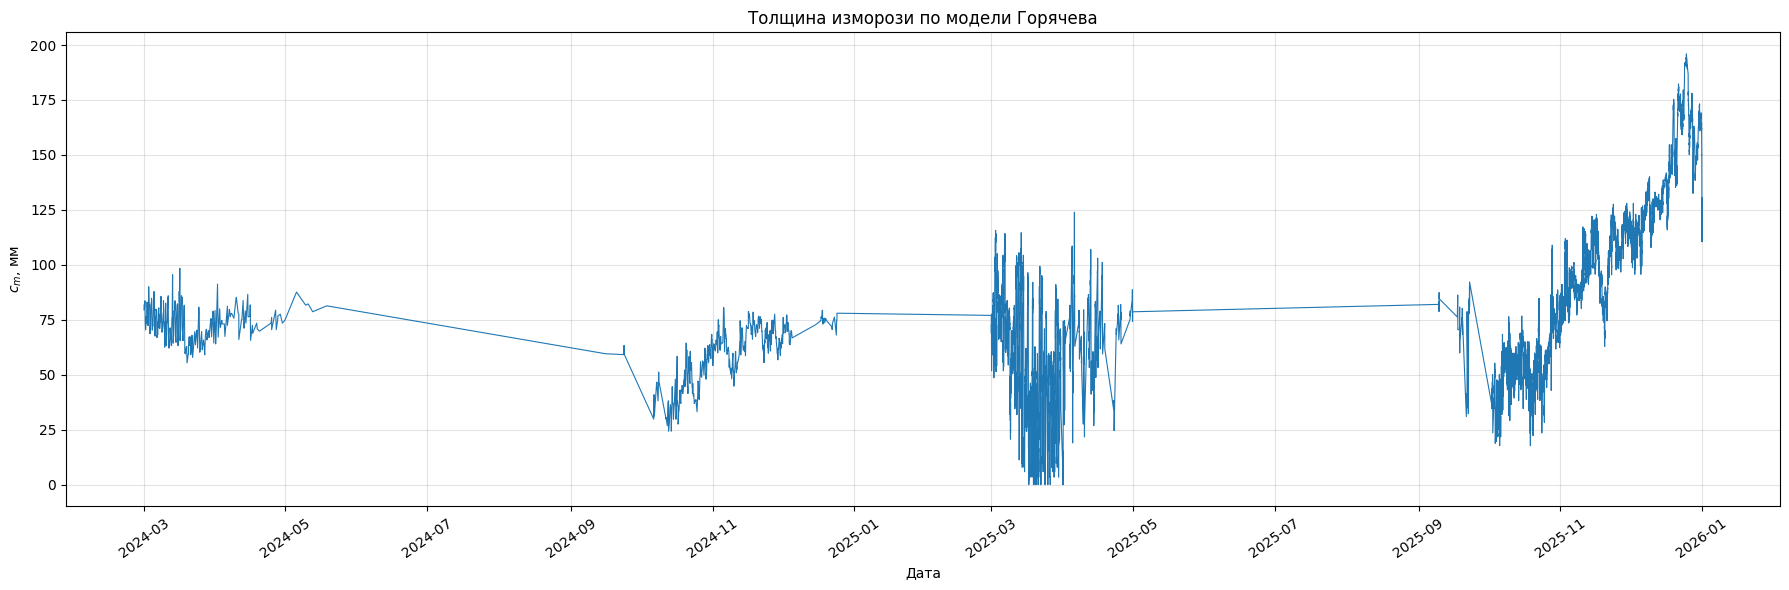

Строк gorStatus = ok: 16108
Максимальная толщина, мм: 195.974
Медианная толщина по valid rows, мм: 86.987


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


df_gor_simple = (
    df_sim[
        [
            "timestamp",
            "gorCm",
            "gorStatus",
        ]
    ]
    .copy()
)

df_gor_simple["timestamp"] = pd.to_datetime(
    df_gor_simple["timestamp"],
    errors="coerce",
)

df_gor_simple["gorCmMm"] = (
    pd.to_numeric(
        df_gor_simple["gorCm"],
        errors="coerce",
    )
    * 1000.0
)

df_gor_simple = (
    df_gor_simple
    .dropna(
        subset=["timestamp"]
    )
    .sort_values("timestamp")
)


gor_ok_mask = (
    df_gor_simple["gorStatus"]
    .eq("ok")
    & df_gor_simple["gorCmMm"].notna()
)


plt.figure(
    figsize=(18, 6)
)

plt.plot(
    df_gor_simple.loc[
        gor_ok_mask,
        "timestamp",
    ],
    df_gor_simple.loc[
        gor_ok_mask,
        "gorCmMm",
    ],
    color="tab:blue",
    linewidth=0.8,
)

plt.title(
    "Толщина изморози по модели Горячева"
)

plt.xlabel(
    "Дата"
)

plt.ylabel(
    "$c_m$, мм"
)

plt.grid(
    True,
    alpha=0.35,
)

plt.gca().xaxis.set_major_locator(
    mdates.MonthLocator(
        interval=2,
    )
)

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter(
        "%Y-%m"
    )
)

plt.xticks(
    rotation=35
)

plt.tight_layout()
plt.show()


print(
    "Строк gorStatus = ok:",
    int(gor_ok_mask.sum()),
)

print(
    "Максимальная толщина, мм:",
    round(
        float(
            df_gor_simple.loc[
                gor_ok_mask,
                "gorCmMm",
            ].max()
        ),
        3,
    ),
)

print(
    "Медианная толщина по valid rows, мм:",
    round(
        float(
            df_gor_simple.loc[
                gor_ok_mask,
                "gorCmMm",
            ].median()
        ),
        3,
    ),
)

In [ ]:
from pathlib import Path
import math

import numpy as np
import pandas as pd

from src.goryachev_model import (
    eq1_q0_from_temperature,
    eq5_L0g,
    eq6_tension,
    eq7_sag,
    eq12_ice_wall_thickness,
)


def resolve_required_column(
    dataframe: pd.DataFrame,
    candidates: list[str],
    semantic_name: str,
) -> str:
    for column in candidates:
        if column in dataframe.columns:
            return column

    related_columns = [
        column
        for column in dataframe.columns
        if any(
            token in column.lower()
            for token in [
                "reference",
                "segment",
                "timestamp",
                "rho",
                "t1",
                "gor",
                "phi",
                "key",
            ]
        )
    ]

    raise KeyError(
        f"Cannot resolve {semantic_name}. "
        f"Candidates: {candidates}. "
        f"Related available columns: "
        f"{related_columns}"
    )


assert "df_goryachev_reference_states" in globals(), (
    "df_goryachev_reference_states is unavailable."
)

assert "df_cal" in globals(), (
    "df_cal is unavailable."
)

assert "df_sim" in globals(), (
    "df_sim is unavailable."
)

assert "cable_params" in globals(), (
    "cable_params is unavailable."
)


SIM_TIMESTAMP_COLUMN = resolve_required_column(
    dataframe=df_sim,
    candidates=[
        "timestamp",
    ],
    semantic_name="simulation timestamp",
)

CAL_TIMESTAMP_COLUMN = resolve_required_column(
    dataframe=df_cal,
    candidates=[
        "timestamp",
    ],
    semantic_name="calibration timestamp",
)

SIM_REFERENCE_KEY_COLUMN = resolve_required_column(
    dataframe=df_sim,
    candidates=[
        "gorReferenceKey",
        "goryachevReferenceKey",
        "orientationReferenceKey",
    ],
    semantic_name="simulation reference key",
)

REFERENCE_KEY_COLUMN = resolve_required_column(
    dataframe=df_goryachev_reference_states,
    candidates=[
        "goryachevReferenceKey",
        "gorReferenceKey",
        "orientationReferenceKey",
    ],
    semantic_name="reference-state key",
)

T1_COLUMN = resolve_required_column(
    dataframe=df_sim,
    candidates=[
        "T1C",
        "t1C",
    ],
    semantic_name="wire temperature",
)

RHO_COLUMN = resolve_required_column(
    dataframe=df_sim,
    candidates=[
        "rhotkgm3",
        "rhoTkgm3",
    ],
    semantic_name="Makkonen density",
)

GOR_STATUS_COLUMN = resolve_required_column(
    dataframe=df_sim,
    candidates=[
        "gorStatus",
    ],
    semantic_name="Goryachev status",
)

GOR_L0G_COLUMN = resolve_required_column(
    dataframe=df_sim,
    candidates=[
        "gorL0gM",
        "gorL0g",
    ],
    semantic_name="current runtime L0g",
)

GOR_FG_COLUMN = resolve_required_column(
    dataframe=df_sim,
    candidates=[
        "gorFgN",
    ],
    semantic_name="current runtime Fg",
)

GOR_SAG_COLUMN = resolve_required_column(
    dataframe=df_sim,
    candidates=[
        "gorSagM",
    ],
    semantic_name="current runtime sag",
)

GOR_CM_COLUMN = resolve_required_column(
    dataframe=df_sim,
    candidates=[
        "gorCm",
    ],
    semantic_name="current runtime thickness",
)

PHI_H_COLUMN = resolve_required_column(
    dataframe=df_cal,
    candidates=[
        "phiHdeg",
    ],
    semantic_name="phiH",
)

PHI_K1_COLUMN = resolve_required_column(
    dataframe=df_cal,
    candidates=[
        "phiK1deg",
    ],
    semantic_name="phiK1",
)


required_reference_columns = [
    REFERENCE_KEY_COLUMN,
    "L0TCalM",
    "phiK0CalDeg",
    "alphaStarPerN",
    "FgCalN",
]

missing_reference_columns = [
    column
    for column in required_reference_columns
    if column not in df_goryachev_reference_states.columns
]

assert not missing_reference_columns, (
    "Reference table is missing columns: "
    f"{missing_reference_columns}"
)


print("L0T-ANCHORED DIAGNOSTIC: RESOLVED COLUMNS")
print("=" * 78)

print("Simulation reference key:", SIM_REFERENCE_KEY_COLUMN)
print("Reference-table key:", REFERENCE_KEY_COLUMN)
print("Wire temperature:", T1_COLUMN)
print("Makkonen density:", RHO_COLUMN)
print("Current runtime L0g:", GOR_L0G_COLUMN)
print("Current runtime Fg:", GOR_FG_COLUMN)
print("Current runtime sag:", GOR_SAG_COLUMN)
print("Current runtime c_m:", GOR_CM_COLUMN)
print("phiH:", PHI_H_COLUMN)
print("phiK1:", PHI_K1_COLUMN)


df_sim_anchor = (
    df_sim[
        [
            SIM_TIMESTAMP_COLUMN,
            SIM_REFERENCE_KEY_COLUMN,
            T1_COLUMN,
            RHO_COLUMN,
            GOR_STATUS_COLUMN,
            GOR_L0G_COLUMN,
            GOR_FG_COLUMN,
            GOR_SAG_COLUMN,
            GOR_CM_COLUMN,
        ]
    ]
    .copy()
    .rename(
        columns={
            SIM_TIMESTAMP_COLUMN: "timestamp",
            SIM_REFERENCE_KEY_COLUMN: "referenceKey",
            T1_COLUMN: "T1C",
            RHO_COLUMN: "rhotkgm3",
            GOR_STATUS_COLUMN: "gorStatus",
            GOR_L0G_COLUMN: "gorL0gCurrentM",
            GOR_FG_COLUMN: "gorFgCurrentN",
            GOR_SAG_COLUMN: "gorSagCurrentM",
            GOR_CM_COLUMN: "gorCmCurrentM",
        }
    )
)

df_cal_anchor = (
    df_cal[
        [
            CAL_TIMESTAMP_COLUMN,
            PHI_H_COLUMN,
            PHI_K1_COLUMN,
        ]
    ]
    .copy()
    .rename(
        columns={
            CAL_TIMESTAMP_COLUMN: "timestamp",
            PHI_H_COLUMN: "phiHdeg",
            PHI_K1_COLUMN: "phiK1deg",
        }
    )
)

df_reference_anchor = (
    df_goryachev_reference_states[
        [
            REFERENCE_KEY_COLUMN,
            "L0TCalM",
            "phiK0CalDeg",
            "alphaStarPerN",
            "FgCalN",
        ]
    ]
    .copy()
    .rename(
        columns={
            REFERENCE_KEY_COLUMN: "referenceKey",
            "L0TCalM": "referenceL0TCalM",
            "phiK0CalDeg": "referencePhiK0CalDeg",
            "alphaStarPerN": "referenceAlphaStarPerN",
            "FgCalN": "referenceFgCalN",
        }
    )
)


for dataframe in [
    df_sim_anchor,
    df_cal_anchor,
]:
    dataframe["timestamp"] = pd.to_datetime(
        dataframe["timestamp"],
        errors="coerce",
    )

    dataframe.dropna(
        subset=["timestamp"],
        inplace=True,
    )

    dataframe.sort_values(
        "timestamp",
        inplace=True,
    )

    dataframe.drop_duplicates(
        subset=["timestamp"],
        keep="last",
        inplace=True,
    )


assert df_sim_anchor["timestamp"].is_unique
assert df_cal_anchor["timestamp"].is_unique
assert df_reference_anchor["referenceKey"].is_unique


df_gor_l0t_anchor = (
    df_sim_anchor
    .merge(
        df_cal_anchor,
        on="timestamp",
        how="left",
        validate="one_to_one",
    )
    .merge(
        df_reference_anchor,
        on="referenceKey",
        how="left",
        validate="many_to_one",
    )
    .sort_values("timestamp")
    .reset_index(drop=True)
)


numeric_columns = [
    "T1C",
    "rhotkgm3",
    "gorL0gCurrentM",
    "gorFgCurrentN",
    "gorSagCurrentM",
    "gorCmCurrentM",
    "phiHdeg",
    "phiK1deg",
    "referenceL0TCalM",
    "referencePhiK0CalDeg",
    "referenceAlphaStarPerN",
    "referenceFgCalN",
]

for column in numeric_columns:
    df_gor_l0t_anchor[column] = pd.to_numeric(
        df_gor_l0t_anchor[column],
        errors="coerce",
    )


df_gor_l0t_anchor["gorStatus"] = (
    df_gor_l0t_anchor["gorStatus"]
    .astype("string")
)


df_gor_l0t_anchor["gorL0gAnchoredM"] = np.nan
df_gor_l0t_anchor["gorFgAnchoredN"] = np.nan
df_gor_l0t_anchor["gorSagAnchoredM"] = np.nan
df_gor_l0t_anchor["gorCmAnchoredM"] = np.nan
df_gor_l0t_anchor["gorDeltaFgAnchoredN"] = np.nan
df_gor_l0t_anchor["gorL0gAnchorStatus"] = (
    "not_calculated"
)


anchored_input_mask = (
    df_gor_l0t_anchor["gorStatus"]
    .eq("ok")
    & df_gor_l0t_anchor["T1C"].notna()
    & df_gor_l0t_anchor["rhotkgm3"].gt(0.0)
    & df_gor_l0t_anchor["phiHdeg"].notna()
    & df_gor_l0t_anchor["phiK1deg"].notna()
    & df_gor_l0t_anchor[
        "referenceL0TCalM"
    ].gt(0.0)
    & df_gor_l0t_anchor[
        "referenceAlphaStarPerN"
    ].gt(0.0)
    & df_gor_l0t_anchor[
        "referencePhiK0CalDeg"
    ].notna()
    & df_gor_l0t_anchor[
        "referenceFgCalN"
    ].notna()
)


for row_index in df_gor_l0t_anchor.index[
    anchored_input_mask
]:
    row = df_gor_l0t_anchor.loc[row_index]

    try:
        q0_now = eq1_q0_from_temperature(
            T1=float(row["T1C"]),
            q0T=float(cable_params.q0TNperm),
            beta=float(cable_params.beta1perC),
            T0=float(cable_params.T0C),
        )

        l0g_anchored = eq5_L0g(
            L0T=float(
                row["referenceL0TCalM"]
            ),
            T1=float(row["T1C"]),
            beta=float(
                cable_params.beta1perC
            ),
            T0=float(cable_params.T0C),
        )

        fg_anchored = eq6_tension(
            phiH_deg=float(row["phiHdeg"]),
            phiK1_rad=math.radians(
                float(row["phiK1deg"])
            ),
            phiK0_rad=math.radians(
                float(
                    row[
                        "referencePhiK0CalDeg"
                    ]
                )
            ),
            alpha_star=float(
                row[
                    "referenceAlphaStarPerN"
                ]
            ),
            L0g=float(l0g_anchored),
            l=float(cable_params.lm),
            B=float(cable_params.BNm2),
            C=float(cable_params.CNm),
        )

        sag_anchored = eq7_sag(
            phiH_deg=float(row["phiHdeg"]),
            L0=float(l0g_anchored),
            alpha_star=float(
                row[
                    "referenceAlphaStarPerN"
                ]
            ),
            q0=float(q0_now),
        )

        if fg_anchored <= 0.0:
            df_gor_l0t_anchor.loc[
                row_index,
                "gorL0gAnchorStatus",
            ] = "anchored_nonpositive_Fg"

            continue

        cm_anchored = eq12_ice_wall_thickness(
            d_pr=float(cable_params.dprm),
            Fg=float(fg_anchored),
            q0g=float(row["rhotkgm3"]),
            L0g=float(l0g_anchored),
        )

        df_gor_l0t_anchor.loc[
            row_index,
            "gorL0gAnchoredM",
        ] = float(l0g_anchored)

        df_gor_l0t_anchor.loc[
            row_index,
            "gorFgAnchoredN",
        ] = float(fg_anchored)

        df_gor_l0t_anchor.loc[
            row_index,
            "gorSagAnchoredM",
        ] = float(sag_anchored)

        df_gor_l0t_anchor.loc[
            row_index,
            "gorCmAnchoredM",
        ] = float(cm_anchored)

        df_gor_l0t_anchor.loc[
            row_index,
            "gorDeltaFgAnchoredN",
        ] = (
            float(fg_anchored)
            - float(
                row["referenceFgCalN"]
            )
        )

        df_gor_l0t_anchor.loc[
            row_index,
            "gorL0gAnchorStatus",
        ] = "ok"

    except Exception as exc:
        df_gor_l0t_anchor.loc[
            row_index,
            "gorL0gAnchorStatus",
        ] = (
            f"error_{type(exc).__name__}"
        )


df_gor_l0t_anchor["gorCmCurrentMm"] = (
    df_gor_l0t_anchor["gorCmCurrentM"]
    * 1000.0
)

df_gor_l0t_anchor["gorCmAnchoredMm"] = (
    df_gor_l0t_anchor["gorCmAnchoredM"]
    * 1000.0
)

df_gor_l0t_anchor["gorL0gDifferenceM"] = (
    df_gor_l0t_anchor["gorL0gAnchoredM"]
    - df_gor_l0t_anchor["gorL0gCurrentM"]
)

df_gor_l0t_anchor["gorFgDifferenceN"] = (
    df_gor_l0t_anchor["gorFgAnchoredN"]
    - df_gor_l0t_anchor["gorFgCurrentN"]
)

df_gor_l0t_anchor["gorSagDifferenceM"] = (
    df_gor_l0t_anchor["gorSagAnchoredM"]
    - df_gor_l0t_anchor["gorSagCurrentM"]
)

df_gor_l0t_anchor["gorCmDifferenceMm"] = (
    df_gor_l0t_anchor["gorCmAnchoredMm"]
    - df_gor_l0t_anchor["gorCmCurrentMm"]
)


STRICT_DIAGNOSTIC_DIR = Path(
    "/content/hoarfrost_project/"
    "output_angle0042_auto_strict_span151"
)

STRICT_DIAGNOSTIC_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

l0t_anchor_output_path = (
    STRICT_DIAGNOSTIC_DIR
    / "goryachev_l0t_anchored_diagnostic.csv"
)

df_gor_l0t_anchor.to_csv(
    l0t_anchor_output_path,
    index=False,
)

assert l0t_anchor_output_path.exists()
assert l0t_anchor_output_path.stat().st_size > 0


anchored_ok_mask = (
    df_gor_l0t_anchor[
        "gorL0gAnchorStatus"
    ]
    .eq("ok")
)


print("L0T-ANCHORED GORYACHEV DIAGNOSTIC")
print("=" * 78)

print(
    "Total rows:",
    len(df_gor_l0t_anchor),
)

print(
    "Current gorStatus = ok rows:",
    int(
        df_gor_l0t_anchor["gorStatus"]
        .eq("ok")
        .sum()
    ),
)

print(
    "Rows valid for anchored diagnostic:",
    int(
        anchored_ok_mask.sum()
    ),
)

print(
    "Saved diagnostic file:",
    l0t_anchor_output_path,
)


print("\nANCHOR STATUS COUNTS")
display(
    df_gor_l0t_anchor[
        "gorL0gAnchorStatus"
    ]
    .value_counts(
        dropna=False,
    )
    .rename("count")
    .to_frame()
)


comparison_columns = [
    "gorL0gCurrentM",
    "gorL0gAnchoredM",
    "gorL0gDifferenceM",
    "gorFgCurrentN",
    "gorFgAnchoredN",
    "gorFgDifferenceN",
    "gorSagCurrentM",
    "gorSagAnchoredM",
    "gorSagDifferenceM",
    "gorCmCurrentMm",
    "gorCmAnchoredMm",
    "gorCmDifferenceMm",
]

comparison_summary = (
    df_gor_l0t_anchor
    .loc[
        anchored_ok_mask,
        comparison_columns,
    ]
    .describe(
        percentiles=[
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99,
        ]
    )
    .T
)

print("\nCURRENT VS L0T-ANCHORED SUMMARY")
display(comparison_summary)


print("\nTOP 20 ABSOLUTE THICKNESS DIFFERENCES")
display(
    df_gor_l0t_anchor
    .loc[
        anchored_ok_mask
    ]
    .assign(
        absThicknessDifferenceMm=lambda frame: (
            frame["gorCmDifferenceMm"]
            .abs()
        )
    )
    .sort_values(
        "absThicknessDifferenceMm",
        ascending=False,
    )
    .head(20)[
        [
            "timestamp",
            "referenceKey",
            "gorStatus",
            "phiHdeg",
            "phiK1deg",
            "gorL0gCurrentM",
            "gorL0gAnchoredM",
            "gorFgCurrentN",
            "gorFgAnchoredN",
            "gorSagCurrentM",
            "gorSagAnchoredM",
            "gorCmCurrentMm",
            "gorCmAnchoredMm",
            "gorCmDifferenceMm",
        ]
    ]
)

ModuleNotFoundError: No module named 'src'

In [ ]:
import inspect

import src.goryachev_model as goryachev_model


print("GORIACHEV MODEL PATH")
print("=" * 78)

print(
    goryachev_model.__file__
)


print("\nEXPORTED FUNCTIONS")
print("=" * 78)

exported_functions = [
    (
        name,
        function,
    )
    for name, function in inspect.getmembers(
        goryachev_model,
        inspect.isfunction,
    )
    if function.__module__
    == goryachev_model.__name__
]

for name, function in exported_functions:
    print(
        f"{name}{inspect.signature(function)}"
    )


print("\nNAMES CONTAINING FORMULA / EQ / L0 / TENSION / SAG")
print("=" * 78)

for name, function in exported_functions:
    name_lower = name.lower()

    if any(
        token in name_lower
        for token in [
            "eq",
            "formula",
            "q0",
            "l0",
            "tension",
            "force",
            "sag",
            "thickness",
            "ice",
        ]
    ):
        print(
            f"{name}{inspect.signature(function)}"
        )

GORIACHEV MODEL PATH
/content/hoarfrost_project/src/goryachev_model.py

EXPORTED FUNCTIONS
_deg_to_rad(angle_deg: 'float') -> 'float'
_rad_to_deg(angle_rad: 'float') -> 'float'
eq10_sensitivity_T(*args, **kwargs) -> 'None'
eq11_total_error(*args, **kwargs) -> 'None'
eq12_ice_wall_thickness(d_pr: 'float', Fg: 'float', q0g: 'float', L0g: 'float') -> 'float'
eq1_q0_from_temperature(T1: 'float', q0T: 'float', beta: 'float', T0: 'float') -> 'float'
eq2_L0(phiH_deg: 'float', l: 'float', q0: 'float', alpha_star: 'float') -> 'float'
eq3_L0T(L0: 'float', T1: 'float', beta: 'float', T0: 'float') -> 'float'
eq4_phiK0(*args, **kwargs)
eq4_phiK0_rad(phiK1_rad: 'float', phiH_deg: 'float', alpha_star: 'float', q0T: 'float', L0T: 'float', l: 'float', B: 'float', C: 'float') -> 'float'
eq5_L0g(L0T: 'float', T1: 'float', beta: 'float', T0: 'float') -> 'float'
eq6_tension(phiH_deg: 'float', phiK1_rad: 'float', phiK0_rad: 'float', alpha_star: 'float', L0g: 'float', l: 'float', B: 'float', C: 'float') -> '

In [ ]:
from pathlib import Path
import math

import numpy as np
import pandas as pd

from src.goryachev_model import (
    eq1_q0_from_temperature,
    eq5_L0g,
    eq6_tension,
    eq7_sag,
    eq12_ice_wall_thickness,
)


def resolve_required_column(
    dataframe: pd.DataFrame,
    candidates: list[str],
    semantic_name: str,
) -> str:
    for column in candidates:
        if column in dataframe.columns:
            return column

    available_columns = dataframe.columns.tolist()

    related_columns = [
        column
        for column in available_columns
        if any(
            token in column.lower()
            for token in [
                "reference",
                "segment",
                "timestamp",
                "rho",
                "t1",
                "gor",
                "phi",
                "key",
                "l0",
                "fg",
                "alpha",
            ]
        )
    ]

    raise KeyError(
        f"Cannot resolve required column: {semantic_name}. "
        f"Candidates: {candidates}. "
        f"Related available columns: {related_columns}"
    )


def get_cable_parameter(
    parameter_object,
    candidates: list[str],
    semantic_name: str,
) -> float:
    for attribute_name in candidates:
        if hasattr(parameter_object, attribute_name):
            value = getattr(
                parameter_object,
                attribute_name,
            )

            if value is not None:
                return float(value)

    raise AttributeError(
        f"Cannot resolve cable parameter: {semantic_name}. "
        f"Candidates: {candidates}. "
        f"Available attributes: "
        f"{sorted(vars(parameter_object).keys())}"
    )


assert "df_goryachev_reference_states" in globals(), (
    "df_goryachev_reference_states is unavailable."
)

assert "df_cal" in globals(), (
    "df_cal is unavailable."
)

assert "df_sim" in globals(), (
    "df_sim is unavailable."
)

assert "cable_params" in globals(), (
    "cable_params is unavailable."
)


SIM_TIMESTAMP_COLUMN = resolve_required_column(
    dataframe=df_sim,
    candidates=[
        "timestamp",
    ],
    semantic_name="simulation timestamp",
)

CAL_TIMESTAMP_COLUMN = resolve_required_column(
    dataframe=df_cal,
    candidates=[
        "timestamp",
    ],
    semantic_name="calibration timestamp",
)

SIM_REFERENCE_KEY_COLUMN = resolve_required_column(
    dataframe=df_sim,
    candidates=[
        "gorReferenceKey",
        "goryachevReferenceKey",
        "orientationReferenceKey",
    ],
    semantic_name="simulation reference key",
)

REFERENCE_KEY_COLUMN = resolve_required_column(
    dataframe=df_goryachev_reference_states,
    candidates=[
        "goryachevReferenceKey",
        "gorReferenceKey",
        "orientationReferenceKey",
    ],
    semantic_name="reference-state key",
)

T1_COLUMN = resolve_required_column(
    dataframe=df_sim,
    candidates=[
        "T1C",
        "t1C",
    ],
    semantic_name="wire temperature",
)

RHO_COLUMN = resolve_required_column(
    dataframe=df_sim,
    candidates=[
        "rhotkgm3",
        "rhoTkgm3",
    ],
    semantic_name="Makkonen ice density",
)

GOR_STATUS_COLUMN = resolve_required_column(
    dataframe=df_sim,
    candidates=[
        "gorStatus",
    ],
    semantic_name="Goryachev status",
)

GOR_L0G_COLUMN = resolve_required_column(
    dataframe=df_sim,
    candidates=[
        "gorL0gM",
        "gorL0g",
    ],
    semantic_name="current runtime L0g",
)

GOR_FG_COLUMN = resolve_required_column(
    dataframe=df_sim,
    candidates=[
        "gorFgN",
    ],
    semantic_name="current runtime Fg",
)

GOR_SAG_COLUMN = resolve_required_column(
    dataframe=df_sim,
    candidates=[
        "gorSagM",
    ],
    semantic_name="current runtime sag",
)

GOR_CM_COLUMN = resolve_required_column(
    dataframe=df_sim,
    candidates=[
        "gorCm",
    ],
    semantic_name="current runtime Goryachev thickness",
)

PHI_H_COLUMN = resolve_required_column(
    dataframe=df_cal,
    candidates=[
        "phiHdeg",
    ],
    semantic_name="phiH angle",
)

PHI_K1_COLUMN = resolve_required_column(
    dataframe=df_cal,
    candidates=[
        "phiK1deg",
    ],
    semantic_name="phiK1 angle",
)

REFERENCE_L0T_COLUMN = resolve_required_column(
    dataframe=df_goryachev_reference_states,
    candidates=[
        "L0TCalM",
        "l0TCalM",
        "referenceL0TCalM",
    ],
    semantic_name="reference L0T",
)

REFERENCE_PHI_K0_COLUMN = resolve_required_column(
    dataframe=df_goryachev_reference_states,
    candidates=[
        "phiK0calRad",
        "phiK0CalRad",
        "phiK0Rad",
        "phiK0rad",
        "phiK0",
        "phiK0calDeg",
        "phiK0CalDeg",
        "phiK0Deg",
        "phiK0deg",
    ],
    semantic_name="reference phiK0",
)

REFERENCE_ALPHA_STAR_COLUMN = resolve_required_column(
    dataframe=df_goryachev_reference_states,
    candidates=[
        "alphaStarPerN",
        "alphaStar1perN",
        "referenceAlphaStarPerN",
    ],
    semantic_name="reference alphaStar",
)

REFERENCE_FG_COLUMN = resolve_required_column(
    dataframe=df_goryachev_reference_states,
    candidates=[
        "FgCalN",
        "fgCalN",
        "referenceFgCalN",
    ],
    semantic_name="reference Fg",
)


REFERENCE_PHI_K0_IS_RAD = (
    "rad"
    in REFERENCE_PHI_K0_COLUMN.lower()
)

REFERENCE_PHI_K0_IS_DEG = (
    "deg"
    in REFERENCE_PHI_K0_COLUMN.lower()
)

assert (
    REFERENCE_PHI_K0_IS_RAD
    or REFERENCE_PHI_K0_IS_DEG
), (
    "Cannot infer units for reference phiK0 from column name: "
    f"{REFERENCE_PHI_K0_COLUMN}. "
    "Expected 'Rad' or 'Deg' in its name."
)


CABLE_Q0T_N_PER_M = get_cable_parameter(
    parameter_object=cable_params,
    candidates=[
        "q0TNperm",
        "q0TNPerM",
        "q0tNperm",
        "q0tNPerM",
    ],
    semantic_name="q0T, N/m",
)

CABLE_BETA_1_PER_C = get_cable_parameter(
    parameter_object=cable_params,
    candidates=[
        "beta1perC",
        "beta1PerC",
    ],
    semantic_name="beta, 1/C",
)

CABLE_T0_C = get_cable_parameter(
    parameter_object=cable_params,
    candidates=[
        "T0C",
        "t0C",
    ],
    semantic_name="T0, C",
)

CABLE_L_M = get_cable_parameter(
    parameter_object=cable_params,
    candidates=[
        "lm",
        "lM",
        "L_M",
    ],
    semantic_name="span length, m",
)

CABLE_B_N_M2 = get_cable_parameter(
    parameter_object=cable_params,
    candidates=[
        "BNm2",
        "bNm2",
        "B_N_M2",
    ],
    semantic_name="B, N*m^2",
)

CABLE_C_N_M = get_cable_parameter(
    parameter_object=cable_params,
    candidates=[
        "CNm",
        "cNm",
        "C_N_M",
    ],
    semantic_name="C, N*m",
)

CABLE_D_PR_M = get_cable_parameter(
    parameter_object=cable_params,
    candidates=[
        "dprm",
        "dPrM",
        "D_PR_M",
    ],
    semantic_name="bare conductor diameter, m",
)


print("L0T-ANCHORED GORYACHEV DIAGNOSTIC")
print("=" * 86)

print(
    "Simulation rows:",
    len(df_sim),
)

print(
    "Calibration rows:",
    len(df_cal),
)

print(
    "Reference-state rows:",
    len(df_goryachev_reference_states),
)

print(
    "Simulation reference key:",
    SIM_REFERENCE_KEY_COLUMN,
)

print(
    "Reference-state key:",
    REFERENCE_KEY_COLUMN,
)

print(
    "Reference L0T:",
    REFERENCE_L0T_COLUMN,
)

print(
    "Reference phiK0:",
    REFERENCE_PHI_K0_COLUMN,
)

print(
    "Reference phiK0 units:",
    "radians"
    if REFERENCE_PHI_K0_IS_RAD
    else "degrees",
)

print(
    "Reference alphaStar:",
    REFERENCE_ALPHA_STAR_COLUMN,
)

print(
    "Reference Fg:",
    REFERENCE_FG_COLUMN,
)


df_sim_anchor = (
    df_sim[
        [
            SIM_TIMESTAMP_COLUMN,
            SIM_REFERENCE_KEY_COLUMN,
            T1_COLUMN,
            RHO_COLUMN,
            GOR_STATUS_COLUMN,
            GOR_L0G_COLUMN,
            GOR_FG_COLUMN,
            GOR_SAG_COLUMN,
            GOR_CM_COLUMN,
        ]
    ]
    .copy()
    .rename(
        columns={
            SIM_TIMESTAMP_COLUMN: "timestamp",
            SIM_REFERENCE_KEY_COLUMN: "referenceKey",
            T1_COLUMN: "T1C",
            RHO_COLUMN: "rhotkgm3",
            GOR_STATUS_COLUMN: "gorStatus",
            GOR_L0G_COLUMN: "gorL0gCurrentM",
            GOR_FG_COLUMN: "gorFgCurrentN",
            GOR_SAG_COLUMN: "gorSagCurrentM",
            GOR_CM_COLUMN: "gorCmCurrentM",
        }
    )
)

df_cal_anchor = (
    df_cal[
        [
            CAL_TIMESTAMP_COLUMN,
            PHI_H_COLUMN,
            PHI_K1_COLUMN,
        ]
    ]
    .copy()
    .rename(
        columns={
            CAL_TIMESTAMP_COLUMN: "timestamp",
            PHI_H_COLUMN: "phiHdeg",
            PHI_K1_COLUMN: "phiK1deg",
        }
    )
)

df_reference_anchor = (
    df_goryachev_reference_states[
        [
            REFERENCE_KEY_COLUMN,
            REFERENCE_L0T_COLUMN,
            REFERENCE_PHI_K0_COLUMN,
            REFERENCE_ALPHA_STAR_COLUMN,
            REFERENCE_FG_COLUMN,
        ]
    ]
    .copy()
    .rename(
        columns={
            REFERENCE_KEY_COLUMN: "referenceKey",
            REFERENCE_L0T_COLUMN: "referenceL0TCalM",
            REFERENCE_PHI_K0_COLUMN: "referencePhiK0Raw",
            REFERENCE_ALPHA_STAR_COLUMN: "referenceAlphaStarPerN",
            REFERENCE_FG_COLUMN: "referenceFgCalN",
        }
    )
)


for dataframe in [
    df_sim_anchor,
    df_cal_anchor,
]:
    dataframe["timestamp"] = pd.to_datetime(
        dataframe["timestamp"],
        errors="coerce",
    )

    dataframe.dropna(
        subset=[
            "timestamp",
        ],
        inplace=True,
    )

    dataframe.sort_values(
        "timestamp",
        inplace=True,
    )

    dataframe.drop_duplicates(
        subset=[
            "timestamp",
        ],
        keep="last",
        inplace=True,
    )


assert df_sim_anchor["timestamp"].is_unique, (
    "df_sim contains duplicate timestamps."
)

assert df_cal_anchor["timestamp"].is_unique, (
    "df_cal contains duplicate timestamps."
)

assert df_reference_anchor["referenceKey"].is_unique, (
    "Reference table contains duplicate reference keys."
)


df_gor_l0t_anchor = (
    df_sim_anchor
    .merge(
        df_cal_anchor,
        on="timestamp",
        how="left",
        validate="one_to_one",
    )
    .merge(
        df_reference_anchor,
        on="referenceKey",
        how="left",
        validate="many_to_one",
    )
    .sort_values(
        "timestamp",
    )
    .reset_index(
        drop=True,
    )
)


numeric_columns = [
    "T1C",
    "rhotkgm3",
    "gorL0gCurrentM",
    "gorFgCurrentN",
    "gorSagCurrentM",
    "gorCmCurrentM",
    "phiHdeg",
    "phiK1deg",
    "referenceL0TCalM",
    "referencePhiK0Raw",
    "referenceAlphaStarPerN",
    "referenceFgCalN",
]

for column in numeric_columns:
    df_gor_l0t_anchor[column] = pd.to_numeric(
        df_gor_l0t_anchor[column],
        errors="coerce",
    )


if REFERENCE_PHI_K0_IS_RAD:
    df_gor_l0t_anchor[
        "referencePhiK0Rad"
    ] = df_gor_l0t_anchor[
        "referencePhiK0Raw"
    ]
else:
    df_gor_l0t_anchor[
        "referencePhiK0Rad"
    ] = np.deg2rad(
        df_gor_l0t_anchor[
            "referencePhiK0Raw"
        ]
    )

df_gor_l0t_anchor[
    "referencePhiK0Deg"
] = np.rad2deg(
    df_gor_l0t_anchor[
        "referencePhiK0Rad"
    ]
)


df_gor_l0t_anchor["gorStatus"] = (
    df_gor_l0t_anchor["gorStatus"]
    .astype("string")
)


df_gor_l0t_anchor["gorL0gAnchoredM"] = np.nan
df_gor_l0t_anchor["gorFgAnchoredN"] = np.nan
df_gor_l0t_anchor["gorSagAnchoredM"] = np.nan
df_gor_l0t_anchor["gorCmAnchoredM"] = np.nan
df_gor_l0t_anchor["gorDeltaFgAnchoredN"] = np.nan
df_gor_l0t_anchor["gorL0gAnchorStatus"] = "not_calculated"


anchored_input_mask = (
    df_gor_l0t_anchor["gorStatus"]
    .eq("ok")
    & df_gor_l0t_anchor["T1C"].notna()
    & df_gor_l0t_anchor["rhotkgm3"].gt(0.0)
    & df_gor_l0t_anchor["phiHdeg"].notna()
    & df_gor_l0t_anchor["phiK1deg"].notna()
    & df_gor_l0t_anchor["referenceL0TCalM"].gt(0.0)
    & df_gor_l0t_anchor[
        "referencePhiK0Rad"
    ].notna()
    & df_gor_l0t_anchor[
        "referenceAlphaStarPerN"
    ].gt(0.0)
    & df_gor_l0t_anchor[
        "referenceFgCalN"
    ].notna()
)


for row_index in df_gor_l0t_anchor.index[
    anchored_input_mask
]:
    row = df_gor_l0t_anchor.loc[
        row_index,
    ]

    try:
        q0_now = eq1_q0_from_temperature(
            T1=float(
                row["T1C"]
            ),
            q0T=CABLE_Q0T_N_PER_M,
            beta=CABLE_BETA_1_PER_C,
            T0=CABLE_T0_C,
        )

        l0g_anchored = eq5_L0g(
            L0T=float(
                row["referenceL0TCalM"]
            ),
            T1=float(
                row["T1C"]
            ),
            beta=CABLE_BETA_1_PER_C,
            T0=CABLE_T0_C,
        )

        fg_anchored = eq6_tension(
            phiH_deg=float(
                row["phiHdeg"]
            ),
            phiK1_rad=math.radians(
                float(
                    row["phiK1deg"]
                )
            ),
            phiK0_rad=float(
                row["referencePhiK0Rad"]
            ),
            alpha_star=float(
                row[
                    "referenceAlphaStarPerN"
                ]
            ),
            L0g=float(
                l0g_anchored
            ),
            l=CABLE_L_M,
            B=CABLE_B_N_M2,
            C=CABLE_C_N_M,
        )

        if (
            not np.isfinite(fg_anchored)
            or fg_anchored <= 0.0
        ):
            df_gor_l0t_anchor.loc[
                row_index,
                "gorL0gAnchorStatus",
            ] = "anchored_nonpositive_or_invalid_Fg"

            continue

        sag_anchored = eq7_sag(
            phiH_deg=float(
                row["phiHdeg"]
            ),
            L0=float(
                l0g_anchored
            ),
            alpha_star=float(
                row[
                    "referenceAlphaStarPerN"
                ]
            ),
            q0=float(
                q0_now
            ),
        )

        cm_anchored = eq12_ice_wall_thickness(
            d_pr=CABLE_D_PR_M,
            Fg=float(
                fg_anchored
            ),
            q0g=float(
                row["rhotkgm3"]
            ),
            L0g=float(
                l0g_anchored
            ),
        )

        if (
            not np.isfinite(cm_anchored)
            or cm_anchored < 0.0
        ):
            df_gor_l0t_anchor.loc[
                row_index,
                "gorL0gAnchorStatus",
            ] = "anchored_invalid_thickness"

            continue

        df_gor_l0t_anchor.loc[
            row_index,
            "gorL0gAnchoredM",
        ] = float(
            l0g_anchored
        )

        df_gor_l0t_anchor.loc[
            row_index,
            "gorFgAnchoredN",
        ] = float(
            fg_anchored
        )

        df_gor_l0t_anchor.loc[
            row_index,
            "gorSagAnchoredM",
        ] = float(
            sag_anchored
        )

        df_gor_l0t_anchor.loc[
            row_index,
            "gorCmAnchoredM",
        ] = float(
            cm_anchored
        )

        df_gor_l0t_anchor.loc[
            row_index,
            "gorDeltaFgAnchoredN",
        ] = (
            float(
                fg_anchored
            )
            - float(
                row[
                    "referenceFgCalN"
                ]
            )
        )

        df_gor_l0t_anchor.loc[
            row_index,
            "gorL0gAnchorStatus",
        ] = "ok"

    except Exception as exc:
        df_gor_l0t_anchor.loc[
            row_index,
            "gorL0gAnchorStatus",
        ] = (
            f"error_{type(exc).__name__}"
        )


df_gor_l0t_anchor["gorCmCurrentMm"] = (
    df_gor_l0t_anchor["gorCmCurrentM"]
    * 1000.0
)

df_gor_l0t_anchor["gorCmAnchoredMm"] = (
    df_gor_l0t_anchor["gorCmAnchoredM"]
    * 1000.0
)

df_gor_l0t_anchor["gorL0gDifferenceM"] = (
    df_gor_l0t_anchor["gorL0gAnchoredM"]
    - df_gor_l0t_anchor["gorL0gCurrentM"]
)

df_gor_l0t_anchor["gorFgDifferenceN"] = (
    df_gor_l0t_anchor["gorFgAnchoredN"]
    - df_gor_l0t_anchor["gorFgCurrentN"]
)

df_gor_l0t_anchor["gorSagDifferenceM"] = (
    df_gor_l0t_anchor["gorSagAnchoredM"]
    - df_gor_l0t_anchor["gorSagCurrentM"]
)

df_gor_l0t_anchor["gorCmDifferenceMm"] = (
    df_gor_l0t_anchor["gorCmAnchoredMm"]
    - df_gor_l0t_anchor["gorCmCurrentMm"]
)


STRICT_DIAGNOSTIC_DIR = Path(
    "/content/hoarfrost_project/"
    "output_angle0042_auto_strict_span151"
)

STRICT_DIAGNOSTIC_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

l0t_anchor_output_path = (
    STRICT_DIAGNOSTIC_DIR
    / "goryachev_l0t_anchored_diagnostic.csv"
)

df_gor_l0t_anchor.to_csv(
    l0t_anchor_output_path,
    index=False,
)

assert l0t_anchor_output_path.exists(), (
    "Diagnostic CSV was not created."
)

assert l0t_anchor_output_path.stat().st_size > 0, (
    "Diagnostic CSV is empty."
)


anchored_ok_mask = (
    df_gor_l0t_anchor[
        "gorL0gAnchorStatus"
    ]
    .eq("ok")
)


print("\nROW COUNTS")
print("=" * 86)

print(
    "Total simulation rows:",
    len(df_gor_l0t_anchor),
)

print(
    "Current gorStatus = ok:",
    int(
        df_gor_l0t_anchor["gorStatus"]
        .eq("ok")
        .sum()
    ),
)

print(
    "Rows with valid L0T-anchored calculation:",
    int(
        anchored_ok_mask.sum()
    ),
)

print(
    "Saved diagnostic CSV:",
    l0t_anchor_output_path,
)


print("\nANCHOR STATUS COUNTS")
print("=" * 86)

display(
    df_gor_l0t_anchor[
        "gorL0gAnchorStatus"
    ]
    .value_counts(
        dropna=False,
    )
    .rename(
        "count"
    )
    .to_frame()
)


print("\nREFERENCE-JOIN CHECK")
print("=" * 86)

reference_join_check = pd.DataFrame(
    {
        "gorStatus_ok_rows": [
            int(
                df_gor_l0t_anchor[
                    "gorStatus"
                ]
                .eq("ok")
                .sum()
            )
        ],
        "missing_reference_L0T": [
            int(
                (
                    df_gor_l0t_anchor[
                        "gorStatus"
                    ]
                    .eq("ok")
                    & df_gor_l0t_anchor[
                        "referenceL0TCalM"
                    ]
                    .isna()
                )
                .sum()
            )
        ],
        "missing_reference_phiK0": [
            int(
                (
                    df_gor_l0t_anchor[
                        "gorStatus"
                    ]
                    .eq("ok")
                    & df_gor_l0t_anchor[
                        "referencePhiK0Rad"
                    ]
                    .isna()
                )
                .sum()
            )
        ],
        "missing_reference_alphaStar": [
            int(
                (
                    df_gor_l0t_anchor[
                        "gorStatus"
                    ]
                    .eq("ok")
                    & df_gor_l0t_anchor[
                        "referenceAlphaStarPerN"
                    ]
                    .isna()
                )
                .sum()
            )
        ],
    }
)

display(
    reference_join_check
)


comparison_columns = [
    "gorL0gCurrentM",
    "gorL0gAnchoredM",
    "gorL0gDifferenceM",
    "gorFgCurrentN",
    "gorFgAnchoredN",
    "gorFgDifferenceN",
    "gorSagCurrentM",
    "gorSagAnchoredM",
    "gorSagDifferenceM",
    "gorCmCurrentMm",
    "gorCmAnchoredMm",
    "gorCmDifferenceMm",
]

comparison_summary = (
    df_gor_l0t_anchor
    .loc[
        anchored_ok_mask,
        comparison_columns,
    ]
    .describe(
        percentiles=[
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99,
        ]
    )
    .T
)

print("\nCURRENT VS L0T-ANCHORED SUMMARY")
print("=" * 86)

display(
    comparison_summary
)


print("\nTOP 20 ABSOLUTE THICKNESS DIFFERENCES")
print("=" * 86)

display(
    df_gor_l0t_anchor
    .loc[
        anchored_ok_mask
    ]
    .assign(
        absThicknessDifferenceMm=lambda frame: (
            frame["gorCmDifferenceMm"]
            .abs()
        )
    )
    .sort_values(
        "absThicknessDifferenceMm",
        ascending=False,
    )
    .head(20)[
        [
            "timestamp",
            "referenceKey",
            "gorStatus",
            "phiHdeg",
            "phiK1deg",
            "referencePhiK0Deg",
            "referenceL0TCalM",
            "gorL0gCurrentM",
            "gorL0gAnchoredM",
            "gorFgCurrentN",
            "gorFgAnchoredN",
            "gorSagCurrentM",
            "gorSagAnchoredM",
            "gorCmCurrentMm",
            "gorCmAnchoredMm",
            "gorCmDifferenceMm",
            "gorL0gAnchorStatus",
        ]
    ]
)

L0T-ANCHORED GORYACHEV DIAGNOSTIC
Simulation rows: 56394
Calibration rows: 56394
Reference-state rows: 16
Simulation reference key: gorReferenceKey
Reference-state key: goryachevReferenceKey
Reference L0T: L0TCalM
Reference phiK0: phiK0calRad
Reference phiK0 units: radians
Reference alphaStar: alphaStarPerN
Reference Fg: FgCalN

ROW COUNTS
Total simulation rows: 56394
Current gorStatus = ok: 15978
Rows with valid L0T-anchored calculation: 15978
Saved diagnostic CSV: /content/hoarfrost_project/output_angle0042_auto_strict_span151/goryachev_l0t_anchored_diagnostic.csv

ANCHOR STATUS COUNTS


,count
gorL0gAnchorStatus,
not_calculated,40416
ok,15978



REFERENCE-JOIN CHECK


,gorStatus_ok_rows,missing_reference_L0T,missing_reference_phiK0,missing_reference_alphaStar
0,15978,0,0,0



CURRENT VS L0T-ANCHORED SUMMARY


,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
gorL0gCurrentM,15978.0,970.872828,28164.532612,1.508358e+02,150.913411,150.932480,150.947132,150.961258,150.977429,150.991013,1.255643e+06
gorL0gAnchoredM,15978.0,150.895327,0.045452,1.508091e+02,150.822466,150.855808,150.901906,150.930028,150.966671,150.979722,1.509922e+02
gorL0gDifferenceM,15978.0,-819.977501,28164.534767,-1.255492e+06,-0.132403,-0.100929,-0.047240,-0.007847,0.039276,0.063537,1.035779e-01
gorFgCurrentN,15978.0,4971.758872,404.472158,8.827176e-01,4482.250350,4716.520660,5015.339559,5218.881020,5386.957696,5578.694411,1.244994e+04
gorFgAnchoredN,15978.0,4997.378693,450.461833,3.001495e+03,4491.188352,4718.923920,5019.768786,5228.668571,5393.197216,5684.396541,1.263799e+04
gorFgDifferenceN,15978.0,25.619821,531.875187,-1.517315e+00,-0.590062,0.125031,0.779502,1.769855,2.313055,2.596410,1.259404e+04
gorSagCurrentM,15978.0,1.905284,9.333656,-1.227386e+00,1.433541,1.585261,1.704025,1.818690,1.961436,2.067080,4.423744e+02
gorSagAnchoredM,15978.0,1.690338,0.322380,-9.715902e+00,1.434132,1.585126,1.703361,1.815946,1.953350,2.066111,5.506325e+00
gorSagDifferenceM,15978.0,-0.214945,9.583597,-4.520903e+02,-0.001659,-0.001188,-0.000542,-0.000084,0.000391,0.000597,8.038762e-04
gorCmCurrentMm,15978.0,140.414750,10.418266,4.034195e-05,132.795739,136.633025,141.324213,144.635167,147.040250,162.861606,2.257644e+02



TOP 20 ABSOLUTE THICKNESS DIFFERENCES


,timestamp,referenceKey,gorStatus,phiHdeg,phiK1deg,referencePhiK0Deg,referenceL0TCalM,gorL0gCurrentM,gorL0gAnchoredM,gorFgCurrentN,gorFgAnchoredN,gorSagCurrentM,gorSagAnchoredM,gorCmCurrentMm,gorCmAnchoredMm,gorCmDifferenceMm,gorL0gAnchorStatus
48666,2025-12-23 19:01:33,3|2025-10,ok,-1.025,13.200,-15.385714,151.00222,86543.111956,150.821887,43.953009,12637.992063,-0.665081,-0.673381,0.028846,227.595336,227.566489,ok
48609,2025-12-23 08:57:22,3|2025-10,ok,-0.945,13.075,-15.385714,151.00222,79777.443007,150.824496,47.465038,12582.415733,-0.615223,-0.620741,0.033779,227.080183,227.046404,ok
48610,2025-12-23 09:08:46,3|2025-10,ok,-0.945,13.075,-15.385714,151.00222,79777.443007,150.824496,47.465038,12582.415733,-0.615223,-0.620741,0.033779,227.080182,227.046403,ok
48611,2025-12-23 09:20:08,3|2025-10,ok,-0.945,13.075,-15.385714,151.00222,79777.443007,150.824496,47.465038,12582.415733,-0.615223,-0.620741,0.033779,227.080180,227.046402,ok
48612,2025-12-23 09:31:34,3|2025-10,ok,-0.945,13.075,-15.385714,151.00222,79777.443007,150.824496,47.465038,12582.415733,-0.615223,-0.620741,0.033779,227.080179,227.046400,ok
48615,2025-12-23 09:54:22,3|2025-10,ok,-0.945,13.075,-15.385714,151.00222,79777.443007,150.824496,47.465038,12582.415733,-0.615223,-0.620741,0.033779,227.080177,227.046398,ok
48614,2025-12-23 09:54:21,3|2025-10,ok,-0.945,13.075,-15.385714,151.00222,79777.443007,150.824496,47.465038,12582.415733,-0.615223,-0.620741,0.033779,227.080177,227.046398,ok
48616,2025-12-23 10:05:44,3|2025-10,ok,-0.945,13.075,-15.385714,151.00222,79777.443007,150.824496,47.465038,12582.415733,-0.615223,-0.620741,0.033779,227.080176,227.046397,ok
48617,2025-12-23 10:17:05,3|2025-10,ok,-0.945,13.075,-15.385714,151.00222,79777.443007,150.824496,47.465038,12582.415733,-0.615223,-0.620741,0.033779,227.080174,227.046396,ok
48619,2025-12-23 10:39:55,3|2025-10,ok,-0.945,13.075,-15.385714,151.00222,79777.443007,150.824496,47.465038,12582.415733,-0.615223,-0.620741,0.033779,227.080172,227.046393,ok


In [ ]:
valid_goryachev_mask = (
    df_gor_l0t_anchor[
        "gorStatus"
    ]
    .eq("ok")
    & df_gor_l0t_anchor[
        "gorL0gCurrentM"
    ]
    .notna()
    & df_gor_l0t_anchor[
        "gorFgCurrentN"
    ]
    .notna()
    & df_gor_l0t_anchor[
        "gorCmCurrentMm"
    ]
    .notna()
)


df_gor_l0t_anchor[
    "isCurrentL0gOutlier"
] = (
    valid_goryachev_mask
    & df_gor_l0t_anchor[
        "gorL0gCurrentM"
    ]
    .gt(200.0)
)


df_gor_l0t_anchor[
    "isCurrentFgLowOutlier"
] = (
    valid_goryachev_mask
    & df_gor_l0t_anchor[
        "gorFgCurrentN"
    ]
    .lt(1000.0)
)


df_gor_l0t_anchor[
    "isCurrentThicknessCollapse"
] = (
    valid_goryachev_mask
    & df_gor_l0t_anchor[
        "gorCmCurrentMm"
    ]
    .lt(1.0)
)


df_gor_l0t_anchor[
    "isRuntimeGoryachevFailure"
] = (
    df_gor_l0t_anchor[
        "isCurrentL0gOutlier"
    ]
    | df_gor_l0t_anchor[
        "isCurrentFgLowOutlier"
    ]
    | df_gor_l0t_anchor[
        "isCurrentThicknessCollapse"
    ]
)


n_valid_goryachev = int(
    valid_goryachev_mask.sum()
)

n_l0g_outliers = int(
    df_gor_l0t_anchor[
        "isCurrentL0gOutlier"
    ]
    .sum()
)

n_fg_outliers = int(
    df_gor_l0t_anchor[
        "isCurrentFgLowOutlier"
    ]
    .sum()
)

n_thickness_collapses = int(
    df_gor_l0t_anchor[
        "isCurrentThicknessCollapse"
    ]
    .sum()
)

n_any_failures = int(
    df_gor_l0t_anchor[
        "isRuntimeGoryachevFailure"
    ]
    .sum()
)


runtime_failure_summary = pd.DataFrame(
    {
        "metric": [
            "Rows in complete simulation table",
            "Current gorStatus = ok rows",
            "Rows valid for failure analysis",
            "Runtime L0g > 200 m",
            "Runtime Fg < 1000 N",
            "Runtime thickness < 1 mm",
            "Any runtime Goryachev failure",
        ],
        "rows": [
            int(
                len(df_gor_l0t_anchor)
            ),
            int(
                df_gor_l0t_anchor[
                    "gorStatus"
                ]
                .eq("ok")
                .sum()
            ),
            n_valid_goryachev,
            n_l0g_outliers,
            n_fg_outliers,
            n_thickness_collapses,
            n_any_failures,
        ],
        "share_of_valid_goryachev_percent": [
            np.nan,
            np.nan,
            100.0,
            100.0
            * n_l0g_outliers
            / n_valid_goryachev,
            100.0
            * n_fg_outliers
            / n_valid_goryachev,
            100.0
            * n_thickness_collapses
            / n_valid_goryachev,
            100.0
            * n_any_failures
            / n_valid_goryachev,
        ],
    }
)


print("CORRECTED RUNTIME GORYACHEV FAILURE SUMMARY")
print("=" * 92)

display(
    runtime_failure_summary
)


runtime_failure_rows = (
    df_gor_l0t_anchor
    .loc[
        df_gor_l0t_anchor[
            "isRuntimeGoryachevFailure"
        ]
    ]
    .copy()
)


runtime_failure_rows[
    "date"
] = runtime_failure_rows[
    "timestamp"
].dt.date


runtime_failure_by_day = (
    runtime_failure_rows
    .groupby(
        "date",
        as_index=False,
    )
    .agg(
        failureRows=(
            "timestamp",
            "size",
        ),
        firstTimestamp=(
            "timestamp",
            "min",
        ),
        lastTimestamp=(
            "timestamp",
            "max",
        ),
        minCurrentL0gM=(
            "gorL0gCurrentM",
            "min",
        ),
        maxCurrentL0gM=(
            "gorL0gCurrentM",
            "max",
        ),
        minCurrentFgN=(
            "gorFgCurrentN",
            "min",
        ),
        maxCurrentFgN=(
            "gorFgCurrentN",
            "max",
        ),
        minAnchoredFgN=(
            "gorFgAnchoredN",
            "min",
        ),
        maxAnchoredFgN=(
            "gorFgAnchoredN",
            "max",
        ),
        minCurrentCmMm=(
            "gorCmCurrentMm",
            "min",
        ),
        maxCurrentCmMm=(
            "gorCmCurrentMm",
            "max",
        ),
        minAnchoredCmMm=(
            "gorCmAnchoredMm",
            "min",
        ),
        maxAnchoredCmMm=(
            "gorCmAnchoredMm",
            "max",
        ),
    )
    .sort_values(
        [
            "date",
            "firstTimestamp",
        ]
    )
    .reset_index(
        drop=True,
    )
)


print("\nVALID RUNTIME FAILURE DAYS ONLY")
print("=" * 92)

display(
    runtime_failure_by_day
)


print("\nALL VALID RUNTIME FAILURE ROWS")
print("=" * 92)

display(
    runtime_failure_rows[
        [
            "timestamp",
            "referenceKey",
            "gorStatus",
            "phiHdeg",
            "phiK1deg",
            "referencePhiK0Deg",
            "referenceL0TCalM",
            "gorL0gCurrentM",
            "gorL0gAnchoredM",
            "gorL0gDifferenceM",
            "gorFgCurrentN",
            "gorFgAnchoredN",
            "gorFgDifferenceN",
            "gorSagCurrentM",
            "gorSagAnchoredM",
            "gorCmCurrentMm",
            "gorCmAnchoredMm",
            "gorCmDifferenceMm",
        ]
    ]
    .sort_values(
        "timestamp",
    )
    .reset_index(
        drop=True,
    )
)


assert (
    runtime_failure_rows[
        "gorStatus"
    ]
    .eq("ok")
    .all()
), (
    "Failure table contains non-valid Goryachev rows."
)

CORRECTED RUNTIME GORYACHEV FAILURE SUMMARY


,metric,rows,share_of_valid_goryachev_percent
0,Rows in complete simulation table,56394,NaN
1,Current gorStatus = ok rows,15978,NaN
2,Rows valid for failure analysis,15978,100.000000
3,Runtime L0g > 200 m,39,0.244086
4,Runtime Fg < 1000 N,39,0.244086
5,Runtime thickness < 1 mm,39,0.244086
6,Any runtime Goryachev failure,39,0.244086



VALID RUNTIME FAILURE DAYS ONLY


,date,failureRows,firstTimestamp,lastTimestamp,minCurrentL0gM,maxCurrentL0gM,minCurrentFgN,maxCurrentFgN,minAnchoredFgN,maxAnchoredFgN,minCurrentCmMm,maxCurrentCmMm,minAnchoredCmMm,maxAnchoredCmMm
0,2025-12-21,1,2025-12-21 02:42:12,2025-12-21 02:42:12,89508.056976,8.950806e+04,17.239741,17.239741,5123.531581,5123.531581,0.010957,0.010957,142.904591,142.904591
1,2025-12-23,32,2025-12-23 04:23:59,2025-12-23 20:32:55,58629.933652,1.253894e+06,0.890832,64.337513,3647.155513,12637.992063,0.000040,0.062147,119.718136,227.595336
2,2025-12-24,6,2025-12-24 03:13:52,2025-12-24 07:24:54,66242.396987,1.255643e+06,0.882718,56.980785,3699.900298,12546.858344,0.000040,0.048772,120.621752,226.753096



ALL VALID RUNTIME FAILURE ROWS


,timestamp,referenceKey,gorStatus,phiHdeg,phiK1deg,referencePhiK0Deg,referenceL0TCalM,gorL0gCurrentM,gorL0gAnchoredM,gorL0gDifferenceM,gorFgCurrentN,gorFgAnchoredN,gorFgDifferenceN,gorSagCurrentM,gorSagAnchoredM,gorCmCurrentMm,gorCmAnchoredMm,gorCmDifferenceMm
0,2025-12-21 02:42:12,3|2025-10,ok,-1.060,-3.790,-15.385714,151.00222,8.950806e+04,150.829135,-8.935723e+04,17.239741,5123.531581,5106.291840,-0.686664,-0.696450,0.010957,142.904591,142.893634
1,2025-12-23 04:23:59,3|2025-10,ok,-14.145,-7.255,-15.385714,151.00222,1.208525e+06,150.824206,-1.208375e+06,0.896699,3647.155513,3646.258815,378.755958,-9.355146,0.000042,119.718136,119.718094
2,2025-12-23 04:35:21,3|2025-10,ok,-14.145,-7.255,-15.385714,151.00222,1.208525e+06,150.824206,-1.208375e+06,0.896699,3647.155513,3646.258815,378.755958,-9.355146,0.000042,119.718136,119.718094
3,2025-12-23 06:40:40,3|2025-10,ok,-1.155,12.895,-15.385714,151.00222,9.754143e+04,150.824206,-9.739061e+04,38.588534,12503.193477,12464.604943,-0.744439,-0.758952,0.022483,226.346881,226.324398
4,2025-12-23 08:45:58,3|2025-10,ok,-0.965,12.865,-15.385714,151.00222,8.146906e+04,150.824206,-8.131824e+04,46.138323,12489.534885,12443.396562,-0.627752,-0.633903,0.032157,226.220164,226.188007
5,2025-12-23 08:57:22,3|2025-10,ok,-0.945,13.075,-15.385714,151.00222,7.977744e+04,150.824496,-7.962662e+04,47.465038,12582.415733,12534.950696,-0.615223,-0.620741,0.033779,227.080183,227.046404
6,2025-12-23 09:08:46,3|2025-10,ok,-0.945,13.075,-15.385714,151.00222,7.977744e+04,150.824496,-7.962662e+04,47.465038,12582.415733,12534.950696,-0.615223,-0.620741,0.033779,227.080182,227.046403
7,2025-12-23 09:20:08,3|2025-10,ok,-0.945,13.075,-15.385714,151.00222,7.977744e+04,150.824496,-7.962662e+04,47.465038,12582.415733,12534.950696,-0.615223,-0.620741,0.033779,227.080180,227.046402
8,2025-12-23 09:31:34,3|2025-10,ok,-0.945,13.075,-15.385714,151.00222,7.977744e+04,150.824496,-7.962662e+04,47.465038,12582.415733,12534.950696,-0.615223,-0.620741,0.033779,227.080179,227.046400
9,2025-12-23 09:42:57,3|2025-10,ok,-0.945,13.075,-15.385714,151.00222,7.977760e+04,150.824786,-7.962677e+04,47.464947,12582.403646,12534.938700,-0.615223,-0.620742,0.033779,227.079843,227.046064


In [ ]:
from src.goryachev_model import (
    eq1_q0_from_temperature,
    eq2_L0,
    eq3_L0T,
    eq5_L0g,
)


failure_examples = (
    df_gor_l0t_anchor
    .loc[
        df_gor_l0t_anchor[
            "isRuntimeGoryachevFailure"
        ]
    ]
    .copy()
    .sort_values(
        "timestamp",
    )
    .reset_index(
        drop=True,
    )
)


reconstruction_rows = []

for _, row in failure_examples.iterrows():
    q0_now = eq1_q0_from_temperature(
        T1=float(
            row["T1C"]
        ),
        q0T=CABLE_Q0T_N_PER_M,
        beta=CABLE_BETA_1_PER_C,
        T0=CABLE_T0_C,
    )

    l0_signed = eq2_L0(
        phiH_deg=float(
            row["phiHdeg"]
        ),
        l=CABLE_L_M,
        q0=q0_now,
        alpha_star=float(
            row[
                "referenceAlphaStarPerN"
            ]
        ),
    )

    l0t_signed = eq3_L0T(
        L0=l0_signed,
        T1=float(
            row["T1C"]
        ),
        beta=CABLE_BETA_1_PER_C,
        T0=CABLE_T0_C,
    )

    l0g_signed = eq5_L0g(
        L0T=l0t_signed,
        T1=float(
            row["T1C"]
        ),
        beta=CABLE_BETA_1_PER_C,
        T0=CABLE_T0_C,
    )

    l0_abs_phi = eq2_L0(
        phiH_deg=abs(
            float(
                row["phiHdeg"]
            )
        ),
        l=CABLE_L_M,
        q0=q0_now,
        alpha_star=float(
            row[
                "referenceAlphaStarPerN"
            ]
        ),
    )

    l0t_abs_phi = eq3_L0T(
        L0=l0_abs_phi,
        T1=float(
            row["T1C"]
        ),
        beta=CABLE_BETA_1_PER_C,
        T0=CABLE_T0_C,
    )

    l0g_abs_phi = eq5_L0g(
        L0T=l0t_abs_phi,
        T1=float(
            row["T1C"]
        ),
        beta=CABLE_BETA_1_PER_C,
        T0=CABLE_T0_C,
    )

    reconstruction_rows.append(
        {
            "timestamp": row["timestamp"],
            "phiHdeg": row["phiHdeg"],
            "T1C": row["T1C"],
            "gorL0gCurrentM": row["gorL0gCurrentM"],
            "eq2Eq3Eq5SignedL0gM": l0g_signed,
            "signedReconstructionErrorM": (
                l0g_signed
                - row["gorL0gCurrentM"]
            ),
            "eq2Eq3Eq5AbsPhiHL0gM": l0g_abs_phi,
            "referenceL0TCalM": row[
                "referenceL0TCalM"
            ],
            "gorL0gAnchoredM": row[
                "gorL0gAnchoredM"
            ],
        }
    )


df_l0g_reconstruction = pd.DataFrame(
    reconstruction_rows
)

df_l0g_reconstruction[
    "absoluteSignedReconstructionErrorM"
] = (
    df_l0g_reconstruction[
        "signedReconstructionErrorM"
    ]
    .abs()
)


print("CURRENT L0G RECONSTRUCTION TEST")
print("=" * 92)

display(
    df_l0g_reconstruction
    .sort_values(
        "absoluteSignedReconstructionErrorM",
        ascending=False,
    )
)


print("\nRECONSTRUCTION ERROR SUMMARY")
print("=" * 92)

display(
    df_l0g_reconstruction[
        [
            "gorL0gCurrentM",
            "eq2Eq3Eq5SignedL0gM",
            "signedReconstructionErrorM",
            "eq2Eq3Eq5AbsPhiHL0gM",
            "gorL0gAnchoredM",
        ]
    ]
    .describe()
)

CURRENT L0G RECONSTRUCTION TEST


,timestamp,phiHdeg,T1C,gorL0gCurrentM,eq2Eq3Eq5SignedL0gM,signedReconstructionErrorM,eq2Eq3Eq5AbsPhiHL0gM,referenceL0TCalM,gorL0gAnchoredM,absoluteSignedReconstructionErrorM
0,2025-12-21 02:42:12,-1.060,-39.7,8.950806e+04,8.950806e+04,0.0,150.755132,151.00222,150.829135,0.0
1,2025-12-23 04:23:59,-14.145,-41.4,1.208525e+06,1.208525e+06,0.0,152.551294,151.00222,150.824206,0.0
2,2025-12-23 04:35:21,-14.145,-41.4,1.208525e+06,1.208525e+06,0.0,152.551294,151.00222,150.824206,0.0
3,2025-12-23 06:40:40,-1.155,-41.4,9.754143e+04,9.754143e+04,0.0,150.777521,151.00222,150.824206,0.0
4,2025-12-23 08:45:58,-0.965,-41.4,8.146906e+04,8.146906e+04,0.0,150.728788,151.00222,150.824206,0.0
5,2025-12-23 08:57:22,-0.945,-41.3,7.977744e+04,7.977744e+04,0.0,150.722627,151.00222,150.824496,0.0
6,2025-12-23 09:08:46,-0.945,-41.3,7.977744e+04,7.977744e+04,0.0,150.722627,151.00222,150.824496,0.0
7,2025-12-23 09:20:08,-0.945,-41.3,7.977744e+04,7.977744e+04,0.0,150.722627,151.00222,150.824496,0.0
8,2025-12-23 09:31:34,-0.945,-41.3,7.977744e+04,7.977744e+04,0.0,150.722627,151.00222,150.824496,0.0
9,2025-12-23 09:42:57,-0.945,-41.2,7.977760e+04,7.977760e+04,0.0,150.722628,151.00222,150.824786,0.0



RECONSTRUCTION ERROR SUMMARY


,gorL0gCurrentM,eq2Eq3Eq5SignedL0gM,signedReconstructionErrorM,eq2Eq3Eq5AbsPhiHL0gM,gorL0gAnchoredM
count,3.900000e+01,3.900000e+01,39.0,39.000000,39.000000
mean,3.360685e+05,3.360685e+05,0.0,151.142272,150.823403
std,4.668925e+05,4.668925e+05,0.0,0.770104,0.002146
min,5.862993e+04,5.862993e+04,0.0,150.617769,150.818987
25%,7.977744e+04,7.977744e+04,0.0,150.722627,150.822322
50%,7.977760e+04,7.977760e+04,0.0,150.722628,150.824496
75%,2.515744e+05,2.515744e+05,0.0,150.977369,150.824496
max,1.255643e+06,1.255643e+06,0.0,152.677345,150.829135


In [ ]:
!grep -RIn \
    --include="*.py" \
    -E "eq2_L0|eq3_L0T|eq5_L0g|gorL0gM|gorFgN|gorCm" \
    /content/hoarfrost_project/src

/content/hoarfrost_project/src/simulation_runner.py:1713:            "gorL0gM": np.nan,
/content/hoarfrost_project/src/simulation_runner.py:1714:            "gorFgN": np.nan,
/content/hoarfrost_project/src/simulation_runner.py:1716:            "gorCm": np.nan,
/content/hoarfrost_project/src/simulation_runner.py:1742:            result["gorCm"] = 0.0
/content/hoarfrost_project/src/simulation_runner.py:1827:            result["gorCm"] = 0.0
/content/hoarfrost_project/src/simulation_runner.py:1868:                "gorL0gM": mechanical.get(
/content/hoarfrost_project/src/simulation_runner.py:1872:                "gorFgN": mechanical.get(
/content/hoarfrost_project/src/simulation_runner.py:1880:                "gorCm": mechanical.get(
/content/hoarfrost_project/src/event_meteo_audit.py:51:    "FgN": "gorFgN",
/content/hoarfrost_project/src/event_meteo_audit.py:53:    "goryachevThicknessM": "gorCm",
/content/hoarfrost_project/src/goryachev_reference.py:25:    eq2_L0,
/content/hoarfrost_proje

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


assert "df_gor_l0t_anchor" in globals(), (
    "df_gor_l0t_anchor is unavailable. "
    "Run the L0T-anchored diagnostic cell first."
)


df_gor_seasonal = (
    df_gor_l0t_anchor
    .copy()
    .sort_values(
        "timestamp"
    )
    .reset_index(
        drop=True
    )
)


df_gor_seasonal["timestamp"] = pd.to_datetime(
    df_gor_seasonal["timestamp"],
    errors="coerce",
)

df_gor_seasonal = (
    df_gor_seasonal
    .dropna(
        subset=[
            "timestamp",
        ]
    )
    .copy()
)


df_gor_seasonal["month"] = (
    df_gor_seasonal["timestamp"]
    .dt.month
)

df_gor_seasonal["year"] = (
    df_gor_seasonal["timestamp"]
    .dt.year
)

df_gor_seasonal["date"] = (
    df_gor_seasonal["timestamp"]
    .dt.date
)


df_gor_seasonal["season"] = np.select(
    [
        df_gor_seasonal["month"].isin(
            [
                11,
                12,
                1,
                2,
            ]
        ),
        df_gor_seasonal["month"].isin(
            [
                6,
                7,
                8,
            ]
        ),
    ],
    [
        "winter_Nov-Feb",
        "summer_Jun-Aug",
    ],
    default="transition_Mar-May_Sep-Oct",
)


df_gor_seasonal["iceRegime"] = np.where(
    df_gor_seasonal["month"].isin(
        [
            11,
            12,
            1,
            2,
        ]
    ),
    "ice_season_Nov-Feb",
    "non_ice_period_Mar-Oct",
)


df_gor_seasonal["isGoryachevOk"] = (
    df_gor_seasonal[
        "gorStatus"
    ]
    .eq("ok")
)


df_gor_seasonal["isCurrentMechanicallyValid"] = (
    df_gor_seasonal[
        "isGoryachevOk"
    ]
    & df_gor_seasonal[
        "gorL0gCurrentM"
    ]
    .gt(0.0)
    & df_gor_seasonal[
        "gorL0gCurrentM"
    ]
    .le(200.0)
    & df_gor_seasonal[
        "gorFgCurrentN"
    ]
    .gt(0.0)
    & df_gor_seasonal[
        "gorCmCurrentMm"
    ]
    .ge(0.0)
)


df_gor_seasonal["isAnchoredMechanicallyValid"] = (
    df_gor_seasonal[
        "gorL0gAnchorStatus"
    ]
    .eq("ok")
    & df_gor_seasonal[
        "gorL0gAnchoredM"
    ]
    .gt(0.0)
    & df_gor_seasonal[
        "gorL0gAnchoredM"
    ]
    .le(200.0)
    & df_gor_seasonal[
        "gorFgAnchoredN"
    ]
    .gt(0.0)
    & df_gor_seasonal[
        "gorCmAnchoredMm"
    ]
    .ge(0.0)
)


def summarize_thickness(
    dataframe: pd.DataFrame,
    thickness_column: str,
    validity_column: str,
    label: str,
) -> pd.DataFrame:
    rows = []

    for season_name in [
        "winter_Nov-Feb",
        "summer_Jun-Aug",
        "transition_Mar-May_Sep-Oct",
    ]:
        season_rows = dataframe.loc[
            dataframe["season"].eq(
                season_name
            )
        ].copy()

        valid_rows = season_rows.loc[
            season_rows[
                validity_column
            ]
        ].copy()

        thickness_mm = valid_rows[
            thickness_column
        ].dropna()

        n_total = len(season_rows)
        n_valid = len(thickness_mm)

        if n_valid == 0:
            rows.append(
                {
                    "modelVariant": label,
                    "season": season_name,
                    "allRows": n_total,
                    "validRows": 0,
                    "coveragePercent": 0.0,
                    "meanMm": np.nan,
                    "stdMm": np.nan,
                    "coefficientVariationPercent": np.nan,
                    "minMm": np.nan,
                    "p05Mm": np.nan,
                    "p25Mm": np.nan,
                    "medianMm": np.nan,
                    "p75Mm": np.nan,
                    "p95Mm": np.nan,
                    "p99Mm": np.nan,
                    "maxMm": np.nan,
                    "iqrMm": np.nan,
                }
            )

            continue

        q05 = thickness_mm.quantile(
            0.05
        )

        q25 = thickness_mm.quantile(
            0.25
        )

        q50 = thickness_mm.quantile(
            0.50
        )

        q75 = thickness_mm.quantile(
            0.75
        )

        q95 = thickness_mm.quantile(
            0.95
        )

        q99 = thickness_mm.quantile(
            0.99
        )

        mean_mm = thickness_mm.mean()
        std_mm = thickness_mm.std()

        rows.append(
            {
                "modelVariant": label,
                "season": season_name,
                "allRows": n_total,
                "validRows": n_valid,
                "coveragePercent": (
                    100.0
                    * n_valid
                    / n_total
                ),
                "meanMm": mean_mm,
                "stdMm": std_mm,
                "coefficientVariationPercent": (
                    100.0
                    * std_mm
                    / mean_mm
                    if mean_mm > 0.0
                    else np.nan
                ),
                "minMm": thickness_mm.min(),
                "p05Mm": q05,
                "p25Mm": q25,
                "medianMm": q50,
                "p75Mm": q75,
                "p95Mm": q95,
                "p99Mm": q99,
                "maxMm": thickness_mm.max(),
                "iqrMm": q75 - q25,
            }
        )

    return pd.DataFrame(
        rows
    )


seasonal_current_summary = summarize_thickness(
    dataframe=df_gor_seasonal,
    thickness_column="gorCmCurrentMm",
    validity_column="isCurrentMechanicallyValid",
    label="current_runtime_filtered",
)

seasonal_anchored_summary = summarize_thickness(
    dataframe=df_gor_seasonal,
    thickness_column="gorCmAnchoredMm",
    validity_column="isAnchoredMechanicallyValid",
    label="L0T_anchored",
)

df_gor_seasonal_summary = pd.concat(
    [
        seasonal_current_summary,
        seasonal_anchored_summary,
    ],
    ignore_index=True,
)


def summarize_temporal_jumps(
    dataframe: pd.DataFrame,
    thickness_column: str,
    validity_column: str,
    label: str,
    max_gap_hours: float = 2.0,
) -> pd.DataFrame:
    rows = []

    for season_name in [
        "winter_Nov-Feb",
        "summer_Jun-Aug",
        "transition_Mar-May_Sep-Oct",
    ]:
        subset = (
            dataframe
            .loc[
                dataframe["season"]
                .eq(season_name)
                & dataframe[
                    validity_column
                ],
                [
                    "timestamp",
                    thickness_column,
                ],
            ]
            .dropna()
            .sort_values(
                "timestamp"
            )
            .copy()
        )

        if len(subset) < 2:
            rows.append(
                {
                    "modelVariant": label,
                    "season": season_name,
                    "nValidRows": len(subset),
                    "nContinuousSteps": 0,
                    "medianAbsStepMm": np.nan,
                    "p95AbsStepMm": np.nan,
                    "p99AbsStepMm": np.nan,
                    "maxAbsStepMm": np.nan,
                    "medianAbsRateMmPerHour": np.nan,
                    "p95AbsRateMmPerHour": np.nan,
                    "maxAbsRateMmPerHour": np.nan,
                }
            )

            continue

        subset["dtHours"] = (
            subset["timestamp"]
            .diff()
            .dt.total_seconds()
            / 3600.0
        )

        subset["deltaMm"] = (
            subset[thickness_column]
            .diff()
        )

        contiguous_steps = (
            subset
            .loc[
                subset["dtHours"].gt(0.0)
                & subset["dtHours"].le(
                    max_gap_hours
                )
            ]
            .copy()
        )

        contiguous_steps["absDeltaMm"] = (
            contiguous_steps[
                "deltaMm"
            ]
            .abs()
        )

        contiguous_steps["absRateMmPerHour"] = (
            contiguous_steps[
                "absDeltaMm"
            ]
            / contiguous_steps[
                "dtHours"
            ]
        )

        if len(contiguous_steps) == 0:
            rows.append(
                {
                    "modelVariant": label,
                    "season": season_name,
                    "nValidRows": len(subset),
                    "nContinuousSteps": 0,
                    "medianAbsStepMm": np.nan,
                    "p95AbsStepMm": np.nan,
                    "p99AbsStepMm": np.nan,
                    "maxAbsStepMm": np.nan,
                    "medianAbsRateMmPerHour": np.nan,
                    "p95AbsRateMmPerHour": np.nan,
                    "maxAbsRateMmPerHour": np.nan,
                }
            )

            continue

        rows.append(
            {
                "modelVariant": label,
                "season": season_name,
                "nValidRows": len(subset),
                "nContinuousSteps": len(
                    contiguous_steps
                ),
                "medianAbsStepMm": (
                    contiguous_steps[
                        "absDeltaMm"
                    ]
                    .median()
                ),
                "p95AbsStepMm": (
                    contiguous_steps[
                        "absDeltaMm"
                    ]
                    .quantile(0.95)
                ),
                "p99AbsStepMm": (
                    contiguous_steps[
                        "absDeltaMm"
                    ]
                    .quantile(0.99)
                ),
                "maxAbsStepMm": (
                    contiguous_steps[
                        "absDeltaMm"
                    ]
                    .max()
                ),
                "medianAbsRateMmPerHour": (
                    contiguous_steps[
                        "absRateMmPerHour"
                    ]
                    .median()
                ),
                "p95AbsRateMmPerHour": (
                    contiguous_steps[
                        "absRateMmPerHour"
                    ]
                    .quantile(0.95)
                ),
                "maxAbsRateMmPerHour": (
                    contiguous_steps[
                        "absRateMmPerHour"
                    ]
                    .max()
                ),
            }
        )

    return pd.DataFrame(
        rows
    )


seasonal_current_jump_summary = summarize_temporal_jumps(
    dataframe=df_gor_seasonal,
    thickness_column="gorCmCurrentMm",
    validity_column="isCurrentMechanicallyValid",
    label="current_runtime_filtered",
)

seasonal_anchored_jump_summary = summarize_temporal_jumps(
    dataframe=df_gor_seasonal,
    thickness_column="gorCmAnchoredMm",
    validity_column="isAnchoredMechanicallyValid",
    label="L0T_anchored",
)

df_gor_seasonal_jump_summary = pd.concat(
    [
        seasonal_current_jump_summary,
        seasonal_anchored_jump_summary,
    ],
    ignore_index=True,
)


monthly_anchored_summary = (
    df_gor_seasonal
    .loc[
        df_gor_seasonal[
            "isAnchoredMechanicallyValid"
        ]
    ]
    .groupby(
        [
            "year",
            "month",
        ],
        as_index=False,
    )
    .agg(
        validRows=(
            "gorCmAnchoredMm",
            "size",
        ),
        meanThicknessMm=(
            "gorCmAnchoredMm",
            "mean",
        ),
        medianThicknessMm=(
            "gorCmAnchoredMm",
            "median",
        ),
        stdThicknessMm=(
            "gorCmAnchoredMm",
            "std",
        ),
        p05ThicknessMm=(
            "gorCmAnchoredMm",
            lambda series: series.quantile(
                0.05
            ),
        ),
        p95ThicknessMm=(
            "gorCmAnchoredMm",
            lambda series: series.quantile(
                0.95
            ),
        ),
        minThicknessMm=(
            "gorCmAnchoredMm",
            "min",
        ),
        maxThicknessMm=(
            "gorCmAnchoredMm",
            "max",
        ),
    )
)

monthly_anchored_summary[
    "coefficientVariationPercent"
] = (
    100.0
    * monthly_anchored_summary[
        "stdThicknessMm"
    ]
    / monthly_anchored_summary[
        "meanThicknessMm"
    ]
)

monthly_anchored_summary[
    "monthStart"
] = pd.to_datetime(
    {
        "year": monthly_anchored_summary[
            "year"
        ],
        "month": monthly_anchored_summary[
            "month"
        ],
        "day": 1,
    }
)


print("GORYACHEV SEASONAL COVERAGE AND THICKNESS STABILITY")
print("=" * 100)

display(
    df_gor_seasonal_summary
    .sort_values(
        [
            "modelVariant",
            "season",
        ]
    )
    .reset_index(
        drop=True
    )
)


print("\nGORYACHEV TEMPORAL STEP-STABILITY")
print("=" * 100)

display(
    df_gor_seasonal_jump_summary
    .sort_values(
        [
            "modelVariant",
            "season",
        ]
    )
    .reset_index(
        drop=True
    )
)


print("\nMONTHLY L0T-ANCHORED THICKNESS SUMMARY")
print("=" * 100)

display(
    monthly_anchored_summary
    .sort_values(
        "monthStart"
    )
    .reset_index(
        drop=True
    )
)


print("\nCURRENT VS ANCHORED DIFFERENCE IN VALID ROWS")
print("=" * 100)

comparison_subset = (
    df_gor_seasonal
    .loc[
        df_gor_seasonal[
            "isCurrentMechanicallyValid"
        ]
        & df_gor_seasonal[
            "isAnchoredMechanicallyValid"
        ]
    ]
    .copy()
)

comparison_subset[
    "absoluteThicknessDifferenceMm"
] = (
    comparison_subset[
        "gorCmDifferenceMm"
    ]
    .abs()
)

seasonal_difference_summary = (
    comparison_subset
    .groupby(
        "season",
        as_index=False,
    )
    .agg(
        rows=(
            "timestamp",
            "size",
        ),
        meanDifferenceMm=(
            "gorCmDifferenceMm",
            "mean",
        ),
        medianDifferenceMm=(
            "gorCmDifferenceMm",
            "median",
        ),
        p95AbsoluteDifferenceMm=(
            "absoluteThicknessDifferenceMm",
            lambda series: series.quantile(
                0.95
            ),
        ),
        p99AbsoluteDifferenceMm=(
            "absoluteThicknessDifferenceMm",
            lambda series: series.quantile(
                0.99
            ),
        ),
        maxAbsoluteDifferenceMm=(
            "absoluteThicknessDifferenceMm",
            "max",
        ),
    )
)

display(
    seasonal_difference_summary
)

GORYACHEV SEASONAL COVERAGE AND THICKNESS STABILITY


,modelVariant,season,allRows,validRows,coveragePercent,meanMm,stdMm,coefficientVariationPercent,minMm,p05Mm,p25Mm,medianMm,p75Mm,p95Mm,p99Mm,maxMm,iqrMm
0,L0T_anchored,summer_Jun-Aug,9093,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,L0T_anchored,transition_Mar-May_Sep-Oct,22723,7901,34.770937,136.712162,7.853434,5.744503,56.071404,131.937570,134.874512,137.001219,140.145451,141.853285,143.908877,199.392206,5.270939
2,L0T_anchored,winter_Nov-Feb,24578,8077,32.862723,145.072194,7.109554,4.900701,108.076963,137.771824,142.897375,144.670722,146.069219,149.666571,176.501675,227.595336,3.171844
3,current_runtime_filtered,summer_Jun-Aug,9093,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,current_runtime_filtered,transition_Mar-May_Sep-Oct,22723,7901,34.770937,136.707832,7.848858,5.741337,56.062115,131.998551,134.871752,136.975429,140.143194,141.836903,143.881156,199.355359,5.271441
5,current_runtime_filtered,winter_Nov-Feb,24578,8038,32.704044,144.739661,5.230399,3.613660,108.010641,137.667226,142.818512,144.593196,145.973480,148.806403,169.796633,225.764369,3.154968



GORYACHEV TEMPORAL STEP-STABILITY


,modelVariant,season,nValidRows,nContinuousSteps,medianAbsStepMm,p95AbsStepMm,p99AbsStepMm,maxAbsStepMm,medianAbsRateMmPerHour,p95AbsRateMmPerHour,maxAbsRateMmPerHour
0,L0T_anchored,summer_Jun-Aug,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,L0T_anchored,transition_Mar-May_Sep-Oct,7901,7541,4.013791e-04,0.936741,6.982534,74.830272,0.001213,3.627073,209.152934
2,L0T_anchored,winter_Nov-Feb,8077,7761,2.247724e-04,0.502828,1.777784,85.064458,0.001214,2.436795,444.547039
3,current_runtime_filtered,summer_Jun-Aug,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,current_runtime_filtered,transition_Mar-May_Sep-Oct,7901,7541,2.837989e-07,0.937230,6.978573,74.821643,0.000002,3.628864,209.128815
5,current_runtime_filtered,winter_Nov-Feb,8038,7721,8.629665e-06,0.466671,1.507965,83.245273,0.000066,2.373654,436.855659



MONTHLY L0T-ANCHORED THICKNESS SUMMARY


,year,month,validRows,meanThicknessMm,medianThicknessMm,stdThicknessMm,p05ThicknessMm,p95ThicknessMm,minThicknessMm,maxThicknessMm,coefficientVariationPercent,monthStart
0,2024,3,183,134.157789,134.041758,1.816787,131.406286,137.459315,130.786272,138.380227,1.354217,2024-03-01
1,2024,4,50,135.851272,135.928336,1.487892,133.552618,138.222103,132.321506,138.592273,1.095236,2024-04-01
2,2024,5,5,136.459552,136.674352,0.699065,135.713390,137.201984,135.700247,137.284241,0.512287,2024-05-01
3,2024,9,4,136.271044,136.406141,0.477537,135.700230,136.652722,135.598386,136.673508,0.350431,2024-09-01
4,2024,10,144,135.731691,135.685027,1.226409,133.592282,137.737366,132.617074,138.447645,0.903554,2024-10-01
5,2024,11,235,135.714391,135.653500,1.106025,133.927208,137.564055,133.062939,139.127471,0.814965,2024-11-01
6,2024,12,155,135.904948,135.725958,1.052661,134.546558,137.522080,132.443496,140.041424,0.774557,2024-12-01
7,2025,1,14,125.290411,127.019735,11.620774,109.788882,138.215048,108.076963,138.432631,9.275071,2025-01-01
8,2025,3,4427,135.581110,135.508395,2.346594,132.205145,138.875499,130.251866,189.828999,1.730767,2025-03-01
9,2025,4,471,133.116933,138.335948,18.763968,91.252865,140.336765,60.111805,193.330624,14.095854,2025-04-01



CURRENT VS ANCHORED DIFFERENCE IN VALID ROWS


,season,rows,meanDifferenceMm,medianDifferenceMm,p95AbsoluteDifferenceMm,p99AbsoluteDifferenceMm,maxAbsoluteDifferenceMm
0,transition_Mar-May_Sep-Oct,7901,0.004330,0.005393,0.044742,0.063304,0.415832
1,winter_Nov-Feb,8038,0.070972,0.075037,0.103373,0.112010,0.138189


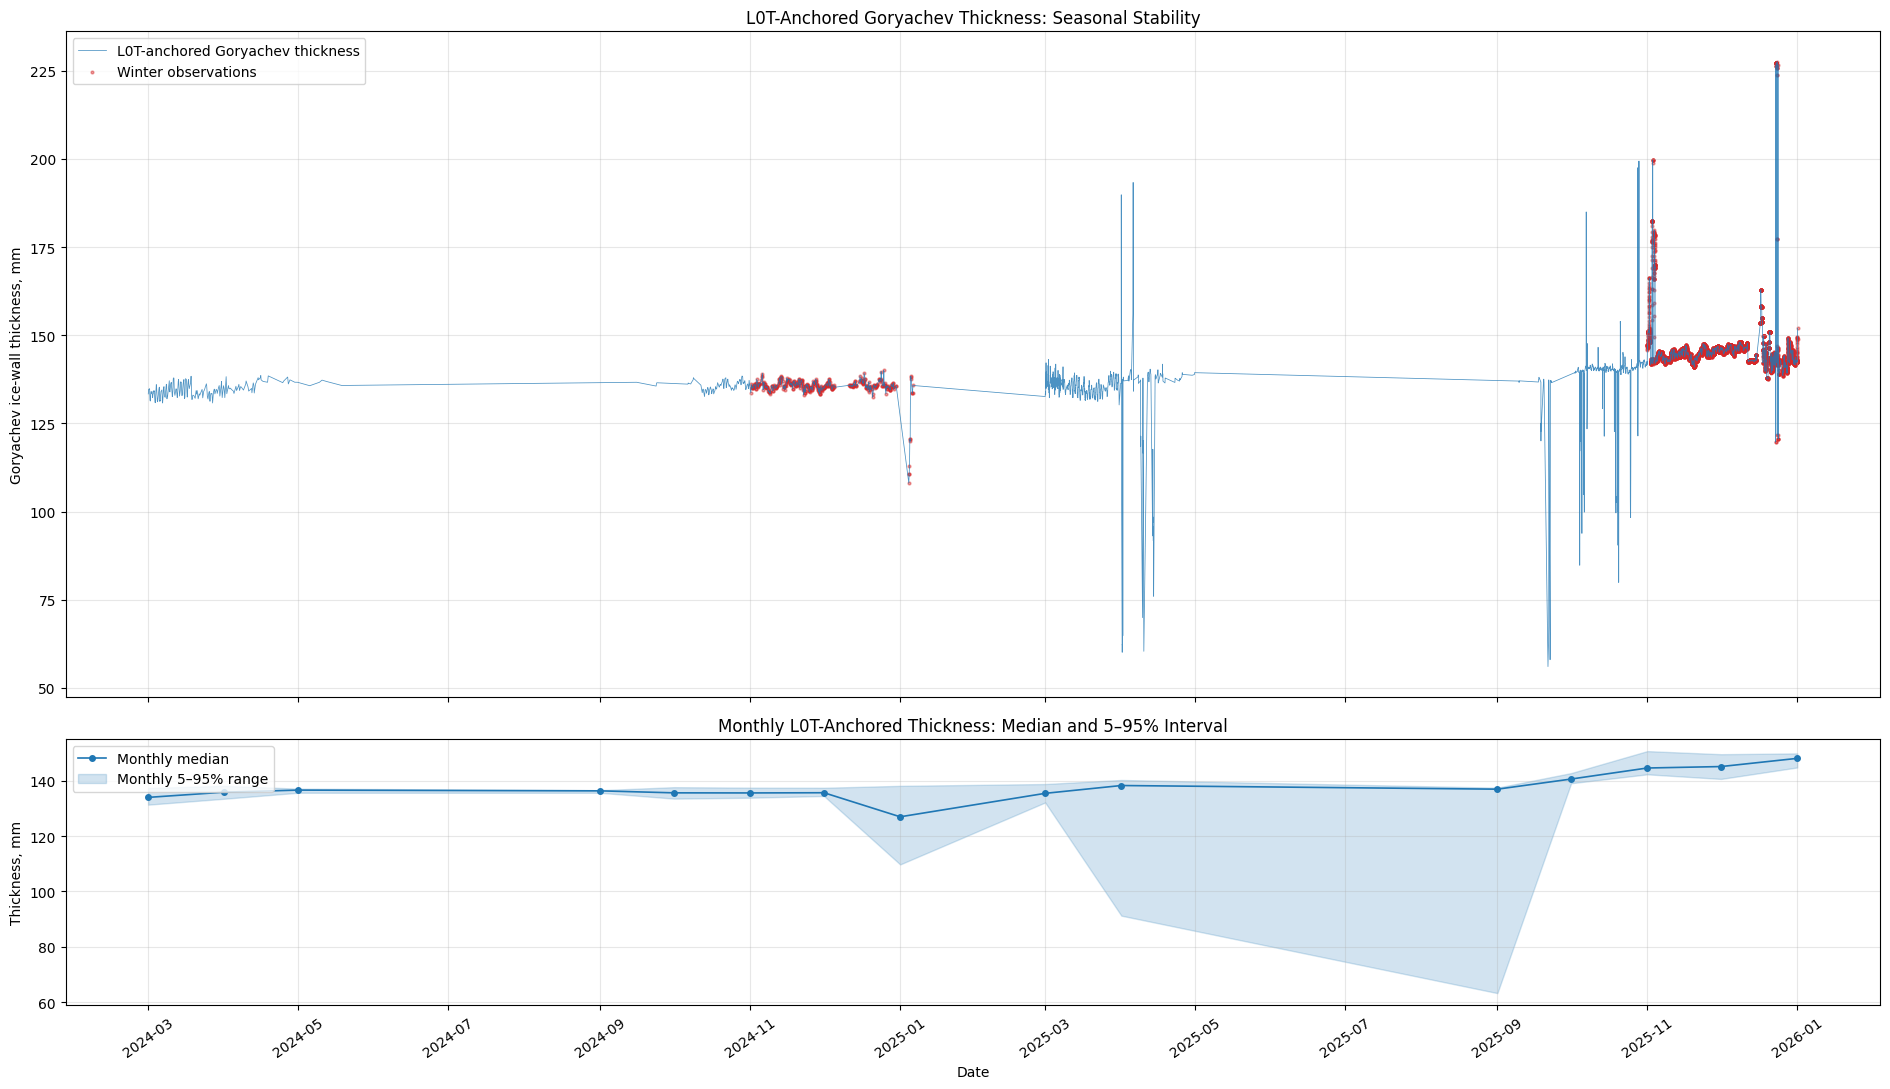

In [ ]:
plot_rows = (
    df_gor_seasonal
    .loc[
        df_gor_seasonal[
            "isAnchoredMechanicallyValid"
        ]
    ]
    .copy()
)


fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(19, 11),
    sharex=True,
    gridspec_kw={
        "height_ratios": [
            2.5,
            1.0,
        ]
    },
)


axes[0].plot(
    plot_rows["timestamp"],
    plot_rows["gorCmAnchoredMm"],
    color="tab:blue",
    linewidth=0.55,
    alpha=0.80,
    label="L0T-anchored Goryachev thickness",
)

axes[0].scatter(
    plot_rows.loc[
        plot_rows[
            "season"
        ]
        .eq("winter_Nov-Feb"),
        "timestamp",
    ],
    plot_rows.loc[
        plot_rows[
            "season"
        ]
        .eq("winter_Nov-Feb"),
        "gorCmAnchoredMm",
    ],
    color="tab:red",
    s=4,
    alpha=0.45,
    label="Winter observations",
)

axes[0].set_title(
    "L0T-Anchored Goryachev Thickness: Seasonal Stability"
)

axes[0].set_ylabel(
    "Goryachev ice-wall thickness, mm"
)

axes[0].grid(
    True,
    alpha=0.3,
)

axes[0].legend(
    loc="upper left",
)


monthly_plot = (
    monthly_anchored_summary
    .sort_values(
        "monthStart"
    )
    .copy()
)

axes[1].plot(
    monthly_plot["monthStart"],
    monthly_plot["medianThicknessMm"],
    color="tab:blue",
    marker="o",
    linewidth=1.2,
    markersize=4,
    label="Monthly median",
)

axes[1].fill_between(
    monthly_plot["monthStart"],
    monthly_plot["p05ThicknessMm"],
    monthly_plot["p95ThicknessMm"],
    color="tab:blue",
    alpha=0.20,
    label="Monthly 5–95% range",
)

axes[1].set_title(
    "Monthly L0T-Anchored Thickness: Median and 5–95% Interval"
)

axes[1].set_xlabel(
    "Date"
)

axes[1].set_ylabel(
    "Thickness, mm"
)

axes[1].grid(
    True,
    alpha=0.3,
)

axes[1].legend(
    loc="upper left",
)


axes[1].xaxis.set_major_locator(
    mdates.MonthLocator(
        interval=2
    )
)

axes[1].xaxis.set_major_formatter(
    mdates.DateFormatter(
        "%Y-%m"
    )
)

plt.xticks(
    rotation=35
)

plt.tight_layout()
plt.show()

In [ ]:
STEP_MAX_GAP_HOURS = 2.0
TOP_N_JUMPS = 30


df_gor_jump_analysis = (
    df_gor_seasonal
    .loc[
        df_gor_seasonal[
            "isAnchoredMechanicallyValid"
        ]
    ]
    .copy()
    .sort_values(
        "timestamp"
    )
    .reset_index(
        drop=True
    )
)


df_gor_jump_analysis[
    "previousTimestamp"
] = df_gor_jump_analysis[
    "timestamp"
].shift(1)

df_gor_jump_analysis[
    "previousThicknessMm"
] = df_gor_jump_analysis[
    "gorCmAnchoredMm"
].shift(1)

df_gor_jump_analysis[
    "previousPhiHdeg"
] = df_gor_jump_analysis[
    "phiHdeg"
].shift(1)

df_gor_jump_analysis[
    "previousPhiK1deg"
] = df_gor_jump_analysis[
    "phiK1deg"
].shift(1)

df_gor_jump_analysis[
    "previousFgN"
] = df_gor_jump_analysis[
    "gorFgAnchoredN"
].shift(1)

df_gor_jump_analysis[
    "previousL0gM"
] = df_gor_jump_analysis[
    "gorL0gAnchoredM"
].shift(1)

df_gor_jump_analysis[
    "previousReferenceKey"
] = df_gor_jump_analysis[
    "referenceKey"
].shift(1)


df_gor_jump_analysis[
    "dtHours"
] = (
    df_gor_jump_analysis[
        "timestamp"
    ]
    - df_gor_jump_analysis[
        "previousTimestamp"
    ]
).dt.total_seconds() / 3600.0


df_gor_jump_analysis[
    "thicknessStepMm"
] = (
    df_gor_jump_analysis[
        "gorCmAnchoredMm"
    ]
    - df_gor_jump_analysis[
        "previousThicknessMm"
    ]
)

df_gor_jump_analysis[
    "absThicknessStepMm"
] = (
    df_gor_jump_analysis[
        "thicknessStepMm"
    ]
    .abs()
)

df_gor_jump_analysis[
    "absThicknessRateMmPerHour"
] = (
    df_gor_jump_analysis[
        "absThicknessStepMm"
    ]
    / df_gor_jump_analysis[
        "dtHours"
    ]
)

df_gor_jump_analysis[
    "phiHStepDeg"
] = (
    df_gor_jump_analysis[
        "phiHdeg"
    ]
    - df_gor_jump_analysis[
        "previousPhiHdeg"
    ]
)

df_gor_jump_analysis[
    "phiK1StepDeg"
] = (
    df_gor_jump_analysis[
        "phiK1deg"
    ]
    - df_gor_jump_analysis[
        "previousPhiK1deg"
    ]
)

df_gor_jump_analysis[
    "FgStepN"
] = (
    df_gor_jump_analysis[
        "gorFgAnchoredN"
    ]
    - df_gor_jump_analysis[
        "previousFgN"
    ]
)

df_gor_jump_analysis[
    "L0gStepM"
] = (
    df_gor_jump_analysis[
        "gorL0gAnchoredM"
    ]
    - df_gor_jump_analysis[
        "previousL0gM"
    ]
)

df_gor_jump_analysis[
    "referenceChanged"
] = (
    df_gor_jump_analysis[
        "referenceKey"
    ]
    .ne(
        df_gor_jump_analysis[
            "previousReferenceKey"
        ]
    )
)


df_gor_jump_analysis = (
    df_gor_jump_analysis
    .loc[
        df_gor_jump_analysis[
            "dtHours"
        ]
        .gt(0.0)
        & df_gor_jump_analysis[
            "dtHours"
        ]
        .le(
            STEP_MAX_GAP_HOURS
        )
    ]
    .copy()
)


top_anchored_jumps = (
    df_gor_jump_analysis
    .sort_values(
        "absThicknessStepMm",
        ascending=False,
    )
    .head(
        TOP_N_JUMPS
    )[
        [
            "timestamp",
            "previousTimestamp",
            "season",
            "iceRegime",
            "dtHours",
            "referenceKey",
            "previousReferenceKey",
            "referenceChanged",
            "previousThicknessMm",
            "gorCmAnchoredMm",
            "thicknessStepMm",
            "absThicknessStepMm",
            "absThicknessRateMmPerHour",
            "previousPhiHdeg",
            "phiHdeg",
            "phiHStepDeg",
            "previousPhiK1deg",
            "phiK1deg",
            "phiK1StepDeg",
            "previousFgN",
            "gorFgAnchoredN",
            "FgStepN",
            "previousL0gM",
            "gorL0gAnchoredM",
            "L0gStepM",
        ]
    ]
)


print("TOP L0T-ANCHORED GORYACHEV THICKNESS JUMPS")
print("=" * 100)

display(
    top_anchored_jumps
)

TOP L0T-ANCHORED GORYACHEV THICKNESS JUMPS


,timestamp,previousTimestamp,season,iceRegime,dtHours,referenceKey,previousReferenceKey,referenceChanged,previousThicknessMm,gorCmAnchoredMm,...,phiHStepDeg,previousPhiK1deg,phiK1deg,phiK1StepDeg,previousFgN,gorFgAnchoredN,FgStepN,previousL0gM,gorL0gAnchoredM,L0gStepM
15126,2025-12-24 04:22:21,2025-12-24 04:10:52,winter_Nov-Feb,ice_season_Nov-Feb,0.191389,3|2025-10,3|2025-10,False,141.688638,226.753096,...,-3.41,-3.985,12.995,16.98,5039.676793,12546.858344,7507.181551,150.821597,150.821887,0.000290
15078,2025-12-23 19:12:57,2025-12-23 19:01:33,winter_Nov-Feb,ice_season_Nov-Feb,0.190000,3|2025-10,3|2025-10,False,227.595336,143.131399,...,3.54,13.200,-3.760,-16.96,12637.992063,5138.960504,-7499.031559,150.821887,150.821307,-0.000580
15127,2025-12-24 04:33:44,2025-12-24 04:22:21,winter_Nov-Feb,ice_season_Nov-Feb,0.189722,3|2025-10,3|2025-10,False,226.753096,142.971063,...,3.31,12.995,-3.785,-16.78,12546.858344,5127.910231,-7418.948113,150.821887,150.822177,0.000290
15012,2025-12-23 06:52:04,2025-12-23 06:40:40,winter_Nov-Feb,ice_season_Nov-Feb,0.190000,3|2025-10,3|2025-10,False,226.346881,142.648996,...,3.67,12.895,-3.835,-16.73,12503.193477,5105.745982,-7397.447495,150.824206,150.824206,0.000000
15043,2025-12-23 13:42:14,2025-12-23 13:19:26,winter_Nov-Feb,ice_season_Nov-Feb,0.380000,3|2025-10,3|2025-10,False,226.343285,142.778274,...,3.47,12.895,-3.815,-16.71,12502.762579,5114.654041,-7388.108538,150.823626,150.823916,0.000290
15011,2025-12-23 06:40:40,2025-12-23 06:17:59,winter_Nov-Feb,ice_season_Nov-Feb,0.378056,3|2025-10,3|2025-10,False,142.843757,226.346881,...,-3.74,-3.805,12.895,16.70,5119.161024,12503.193477,7384.032453,150.823626,150.824206,0.000580
15057,2025-12-23 15:47:52,2025-12-23 15:36:26,winter_Nov-Feb,ice_season_Nov-Feb,0.190556,3|2025-10,3|2025-10,False,142.521247,225.816907,...,0.01,-3.855,12.755,16.61,5096.955996,12446.143289,7349.187293,150.824496,150.824496,0.000000
15023,2025-12-23 08:45:58,2025-12-23 08:34:32,winter_Nov-Feb,ice_season_Nov-Feb,0.190556,3|2025-10,3|2025-10,False,143.035175,226.220164,...,-3.55,-3.775,12.865,16.64,5132.412673,12489.534885,7357.122212,150.824496,150.824206,-0.000290
15061,2025-12-23 16:33:28,2025-12-23 16:22:04,winter_Nov-Feb,ice_season_Nov-Feb,0.190000,3|2025-10,3|2025-10,False,225.734360,142.842261,...,0.00,12.735,-3.805,-16.54,12437.216973,5119.061227,-7318.155746,150.823916,150.823626,-0.000290
15055,2025-12-23 15:36:25,2025-12-23 15:25:03,winter_Nov-Feb,ice_season_Nov-Feb,0.189444,3|2025-10,3|2025-10,False,223.734941,142.521247,...,4.73,12.255,-3.855,-16.11,12223.164972,5096.955996,-7126.208977,150.824496,150.824496,0.000000


WINTER GORYACHEV SEASONAL TRAJECTORY


,iceSeason,dailyPoints,firstDate,lastDate,firstDailyMedianMm,lastDailyMedianMm,netChangeMm,linearTrendMmPerDay,linearTrendMmPer30Days
0,2024/2025,58,2024-11-01,2025-01-06,135.132203,134.726471,-0.405731,-0.043412,-1.302365
1,2025/2026,62,2025-11-01,2026-01-01,150.860706,148.159462,-2.701243,-0.042569,-1.277068



WINTER GORYACHEV MONTHLY ROBUST SUMMARY


,iceSeasonStartYear,monthStart,validRows,meanMm,medianMm,stdMm,p05Mm,p95Mm,minMm,maxMm,monthName,coefficientVariationPercent
0,2024,2024-11-01,235,135.714391,135.653500,1.106025,133.927208,137.564055,133.062939,139.127471,2024-11,0.814965
1,2024,2024-12-01,155,135.904948,135.725958,1.052661,134.546558,137.522080,132.443496,140.041424,2024-12,0.774557
2,2024,2025-01-01,14,125.290411,127.019735,11.620774,109.788882,138.215048,108.076963,138.432631,2025-01,9.275071
3,2025,2025-11-01,4198,145.564625,144.672666,5.444756,142.383742,150.784487,140.986500,199.657610,2025-11,3.740439
4,2025,2025-12-01,3458,145.588714,145.195593,8.338427,140.721409,149.666796,119.718136,227.595336,2025-12,5.727385
5,2025,2026-01-01,17,147.637014,148.159462,2.167736,144.862951,149.957105,144.106167,151.990091,2026-01,1.468288


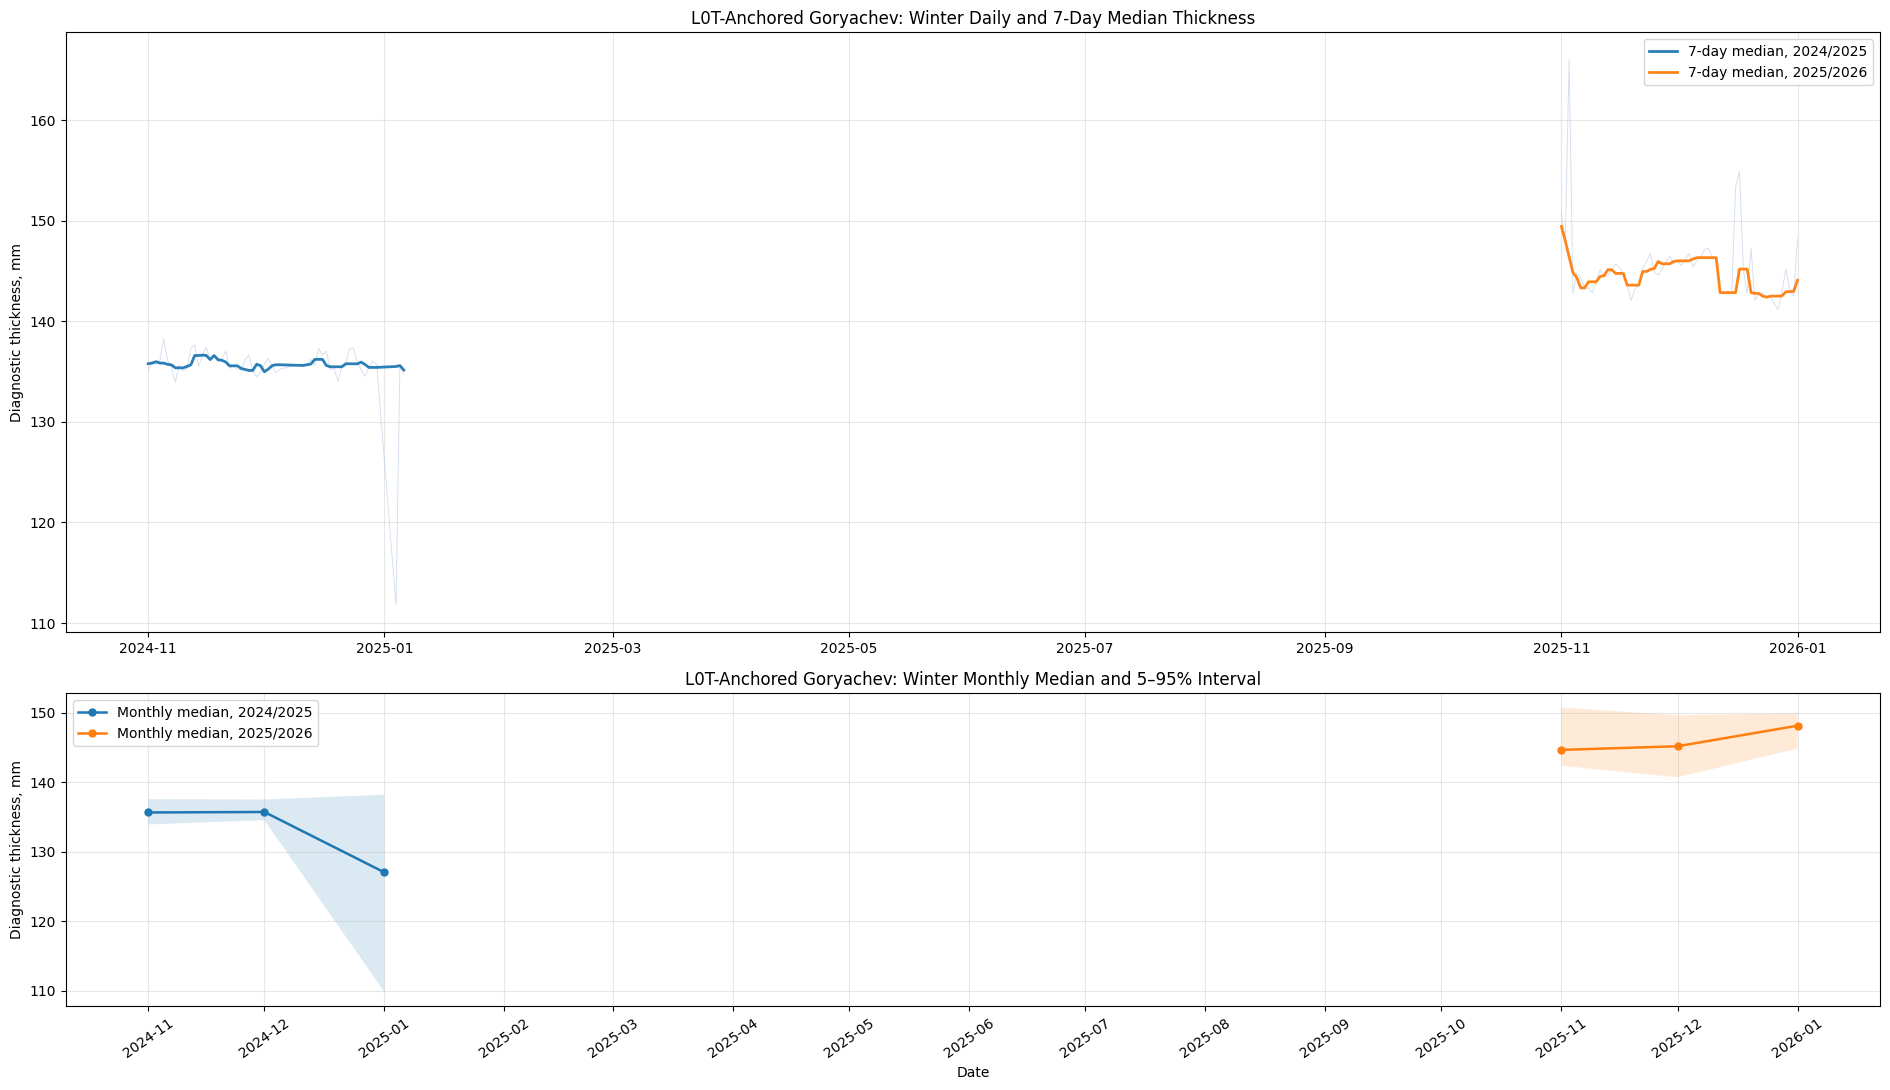

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


assert "df_gor_seasonal" in globals(), (
    "df_gor_seasonal is unavailable. "
    "Run the seasonal L0T-anchored Goryachev diagnostic first."
)


df_gor_season_curve = (
    df_gor_seasonal
    .loc[
        df_gor_seasonal[
            "isAnchoredMechanicallyValid"
        ]
    ]
    .copy()
)


df_gor_season_curve["timestamp"] = pd.to_datetime(
    df_gor_season_curve["timestamp"],
    errors="coerce",
)

df_gor_season_curve = (
    df_gor_season_curve
    .dropna(
        subset=[
            "timestamp",
            "gorCmAnchoredMm",
        ]
    )
    .sort_values(
        "timestamp",
    )
    .reset_index(
        drop=True,
    )
)


df_gor_season_curve["month"] = (
    df_gor_season_curve["timestamp"]
    .dt.month
)

df_gor_season_curve["date"] = (
    df_gor_season_curve["timestamp"]
    .dt.floor(
        "D"
    )
)

df_gor_season_curve["isIceSeason"] = (
    df_gor_season_curve["month"]
    .isin(
        [
            11,
            12,
            1,
            2,
        ]
    )
)

df_gor_season_curve["iceSeasonStartYear"] = np.where(
    df_gor_season_curve["month"].ge(11),
    df_gor_season_curve["timestamp"].dt.year,
    df_gor_season_curve["timestamp"].dt.year - 1,
)


df_gor_winter_curve = (
    df_gor_season_curve
    .loc[
        df_gor_season_curve[
            "isIceSeason"
        ]
    ]
    .copy()
)


daily_goryachev_curve = (
    df_gor_winter_curve
    .groupby(
        [
            "iceSeasonStartYear",
            "date",
        ],
        as_index=False,
    )
    .agg(
        validRows=(
            "gorCmAnchoredMm",
            "size",
        ),
        meanMm=(
            "gorCmAnchoredMm",
            "mean",
        ),
        medianMm=(
            "gorCmAnchoredMm",
            "median",
        ),
        p05Mm=(
            "gorCmAnchoredMm",
            lambda series: series.quantile(
                0.05
            ),
        ),
        p25Mm=(
            "gorCmAnchoredMm",
            lambda series: series.quantile(
                0.25
            ),
        ),
        p75Mm=(
            "gorCmAnchoredMm",
            lambda series: series.quantile(
                0.75
            ),
        ),
        p95Mm=(
            "gorCmAnchoredMm",
            lambda series: series.quantile(
                0.95
            ),
        ),
        minMm=(
            "gorCmAnchoredMm",
            "min",
        ),
        maxMm=(
            "gorCmAnchoredMm",
            "max",
        ),
    )
    .sort_values(
        [
            "iceSeasonStartYear",
            "date",
        ]
    )
    .reset_index(
        drop=True,
    )
)


daily_goryachev_curve[
    "seasonDay"
] = (
    daily_goryachev_curve["date"]
    - pd.to_datetime(
        daily_goryachev_curve[
            "iceSeasonStartYear"
        ]
        .astype(str)
        + "-11-01"
    )
).dt.days + 1


daily_goryachev_curve[
    "rollingMedian7Dmm"
] = (
    daily_goryachev_curve
    .groupby(
        "iceSeasonStartYear"
    )[
        "medianMm"
    ]
    .transform(
        lambda series: (
            series
            .rolling(
                window=7,
                min_periods=3,
                center=True,
            )
            .median()
        )
    )
)


daily_goryachev_curve[
    "rollingMean7Dmm"
] = (
    daily_goryachev_curve
    .groupby(
        "iceSeasonStartYear"
    )[
        "meanMm"
    ]
    .transform(
        lambda series: (
            series
            .rolling(
                window=7,
                min_periods=3,
                center=True,
            )
            .mean()
        )
    )
)


df_gor_winter_monthly = (
    df_gor_winter_curve
    .assign(
        monthStart=lambda frame: (
            frame["timestamp"]
            .dt.to_period("M")
            .dt.to_timestamp()
        )
    )
    .groupby(
        [
            "iceSeasonStartYear",
            "monthStart",
        ],
        as_index=False,
    )
    .agg(
        validRows=(
            "gorCmAnchoredMm",
            "size",
        ),
        meanMm=(
            "gorCmAnchoredMm",
            "mean",
        ),
        medianMm=(
            "gorCmAnchoredMm",
            "median",
        ),
        stdMm=(
            "gorCmAnchoredMm",
            "std",
        ),
        p05Mm=(
            "gorCmAnchoredMm",
            lambda series: series.quantile(
                0.05
            ),
        ),
        p95Mm=(
            "gorCmAnchoredMm",
            lambda series: series.quantile(
                0.95
            ),
        ),
        minMm=(
            "gorCmAnchoredMm",
            "min",
        ),
        maxMm=(
            "gorCmAnchoredMm",
            "max",
        ),
    )
)


df_gor_winter_monthly[
    "monthName"
] = (
    df_gor_winter_monthly[
        "monthStart"
    ]
    .dt.strftime(
        "%Y-%m"
    )
)

df_gor_winter_monthly[
    "coefficientVariationPercent"
] = (
    100.0
    * df_gor_winter_monthly[
        "stdMm"
    ]
    / df_gor_winter_monthly[
        "meanMm"
    ]
)


winter_trend_rows = []

for ice_season_year, group in daily_goryachev_curve.groupby(
    "iceSeasonStartYear"
):
    trend_group = (
        group
        .dropna(
            subset=[
                "medianMm",
                "seasonDay",
            ]
        )
        .copy()
    )

    if len(trend_group) < 7:
        winter_trend_rows.append(
            {
                "iceSeason": (
                    f"{ice_season_year}/"
                    f"{ice_season_year + 1}"
                ),
                "dailyPoints": len(
                    trend_group
                ),
                "firstDate": (
                    trend_group["date"].min()
                    if len(trend_group) > 0
                    else pd.NaT
                ),
                "lastDate": (
                    trend_group["date"].max()
                    if len(trend_group) > 0
                    else pd.NaT
                ),
                "firstDailyMedianMm": np.nan,
                "lastDailyMedianMm": np.nan,
                "netChangeMm": np.nan,
                "linearTrendMmPerDay": np.nan,
                "linearTrendMmPer30Days": np.nan,
            }
        )

        continue

    slope_mm_per_day, intercept = np.polyfit(
        trend_group["seasonDay"],
        trend_group["medianMm"],
        deg=1,
    )

    winter_trend_rows.append(
        {
            "iceSeason": (
                f"{ice_season_year}/"
                f"{ice_season_year + 1}"
            ),
            "dailyPoints": len(
                trend_group
            ),
            "firstDate": trend_group[
                "date"
            ].min(),
            "lastDate": trend_group[
                "date"
            ].max(),
            "firstDailyMedianMm": trend_group[
                "medianMm"
            ].iloc[0],
            "lastDailyMedianMm": trend_group[
                "medianMm"
            ].iloc[-1],
            "netChangeMm": (
                trend_group[
                    "medianMm"
                ].iloc[-1]
                - trend_group[
                    "medianMm"
                ].iloc[0]
            ),
            "linearTrendMmPerDay": (
                slope_mm_per_day
            ),
            "linearTrendMmPer30Days": (
                30.0
                * slope_mm_per_day
            ),
        }
    )


df_gor_winter_trend = pd.DataFrame(
    winter_trend_rows
)


print("WINTER GORYACHEV SEASONAL TRAJECTORY")
print("=" * 100)

display(
    df_gor_winter_trend
    .sort_values(
        "iceSeason"
    )
    .reset_index(
        drop=True
    )
)


print("\nWINTER GORYACHEV MONTHLY ROBUST SUMMARY")
print("=" * 100)

display(
    df_gor_winter_monthly
    .sort_values(
        [
            "iceSeasonStartYear",
            "monthStart",
        ]
    )
    .reset_index(
        drop=True
    )
)


fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(19, 11),
    gridspec_kw={
        "height_ratios": [
            2.3,
            1.2,
        ]
    },
)


for ice_season_year, group in daily_goryachev_curve.groupby(
    "iceSeasonStartYear"
):
    axes[0].plot(
        group["date"],
        group["medianMm"],
        color="lightsteelblue",
        linewidth=0.65,
        alpha=0.55,
    )

    axes[0].plot(
        group["date"],
        group["rollingMedian7Dmm"],
        linewidth=2.0,
        alpha=0.95,
        label=(
            f"7-day median, "
            f"{ice_season_year}/"
            f"{ice_season_year + 1}"
        ),
    )


axes[0].set_title(
    "L0T-Anchored Goryachev: Winter Daily and 7-Day Median Thickness"
)

axes[0].set_ylabel(
    "Diagnostic thickness, mm"
)

axes[0].grid(
    True,
    alpha=0.30,
)

axes[0].legend(
    loc="best"
)


for ice_season_year, group in df_gor_winter_monthly.groupby(
    "iceSeasonStartYear"
):
    axes[1].plot(
        group["monthStart"],
        group["medianMm"],
        marker="o",
        linewidth=1.8,
        markersize=5,
        label=(
            f"Monthly median, "
            f"{ice_season_year}/"
            f"{ice_season_year + 1}"
        ),
    )

    axes[1].fill_between(
        group["monthStart"],
        group["p05Mm"],
        group["p95Mm"],
        alpha=0.16,
    )


axes[1].set_title(
    "L0T-Anchored Goryachev: Winter Monthly Median and 5–95% Interval"
)

axes[1].set_xlabel(
    "Date"
)

axes[1].set_ylabel(
    "Diagnostic thickness, mm"
)

axes[1].grid(
    True,
    alpha=0.30,
)

axes[1].legend(
    loc="best"
)

axes[1].xaxis.set_major_locator(
    mdates.MonthLocator(
        interval=1
    )
)

axes[1].xaxis.set_major_formatter(
    mdates.DateFormatter(
        "%Y-%m"
    )
)

plt.xticks(
    rotation=35
)

plt.tight_layout()
plt.show()

GORYACHEV WINTER DRIVER TRENDS


,iceSeason,variable,dailyPoints,firstDailyMedian,lastDailyMedian,netChange,trendPerDay,trendPer30Days,coefficientVariationPercent
0,2024/2025,gorCmAnchoredMm,58,135.132203,134.726471,-4.057312e-01,-4.341218e-02,-1.302365e+00,2.422828e+00
1,2024/2025,gorFgAnchoredN,58,4604.742011,4577.084743,-2.765727e+01,-2.675780e+00,-8.027339e+01,4.304587e+00
2,2024/2025,gorL0gAnchoredM,58,150.912760,150.866947,-4.581230e-02,-9.324913e-04,-2.797474e-02,1.488911e-02
3,2024/2025,gorMechanicalIndex,58,0.610255,0.606771,-3.484191e-03,-3.508951e-04,-1.052685e-02,4.303251e+00
4,2024/2025,phiHdeg,58,2.445000,2.640000,1.950000e-01,-1.234389e-03,-3.703168e-02,5.402273e+00
5,2024/2025,phiK1deg,58,-3.890000,-3.955000,-6.500000e-02,-6.080713e-03,-1.824214e-01,1.171508e+01
6,2024/2025,rhotkgm3,58,49.999999,49.999998,-8.484580e-07,-7.077209e-09,-2.123163e-07,8.118545e-07
7,2025/2026,gorCmAnchoredMm,62,150.860706,148.159462,-2.701243e+00,-4.256894e-02,-1.277068e+00,2.523763e+00
8,2025/2026,gorFgAnchoredN,62,5077.950668,5493.461070,4.155104e+02,1.096864e+00,3.290592e+01,3.276988e+00
9,2025/2026,gorL0gAnchoredM,62,150.905965,150.844501,-6.146394e-02,-1.338239e-03,-4.014718e-02,1.781216e-02



GORYACHEV THICKNESS-DRIVER SPEARMAN CORRELATIONS


,iceSeason,response,predictor,spearmanCorrelation
0,2024/2025,gorCmAnchoredMm,gorMechanicalIndex,0.999938
1,2024/2025,gorCmAnchoredMm,gorFgAnchoredN,0.999385
2,2024/2025,gorCmAnchoredMm,phiK1deg,0.999031
3,2024/2025,gorCmAnchoredMm,phiHdeg,0.231365
4,2024/2025,gorCmAnchoredMm,rhotkgm3,0.040081
5,2024/2025,gorCmAnchoredMm,gorL0gAnchoredM,-0.154490
6,2025/2026,gorCmAnchoredMm,gorMechanicalIndex,1.000000
7,2025/2026,gorCmAnchoredMm,phiK1deg,0.809144
8,2025/2026,gorCmAnchoredMm,gorFgAnchoredN,0.809071
9,2025/2026,gorCmAnchoredMm,phiHdeg,0.266215



MONTHLY GORYACHEV DRIVER MEDIANS


,iceSeasonStartYear,monthStart,validRows,gorCmAnchoredMm,gorFgAnchoredN,gorL0gAnchoredM,rhotkgm3,phiHdeg,phiK1deg,gorMechanicalIndex
0,2024,2024-11-01,235,135.653500,4638.331146,150.899712,49.999998,2.555,-3.815,0.614788
1,2024,2024-12-01,155,135.725958,4642.901185,150.869847,49.999998,2.545,-3.805,0.615419
2,2024,2025-01-01,14,127.019735,4097.062909,150.857524,49.999998,2.435,-5.040,0.543174
3,2025,2025-11-01,4198,144.672666,5216.097528,150.874073,49.964007,2.685,-3.585,0.695877
4,2025,2025-12-01,3458,145.195593,5282.983096,150.828265,49.984753,2.640,-3.435,0.700732
5,2025,2026-01-01,17,148.159462,5493.461070,150.844501,49.985695,1.945,-2.955,0.728569


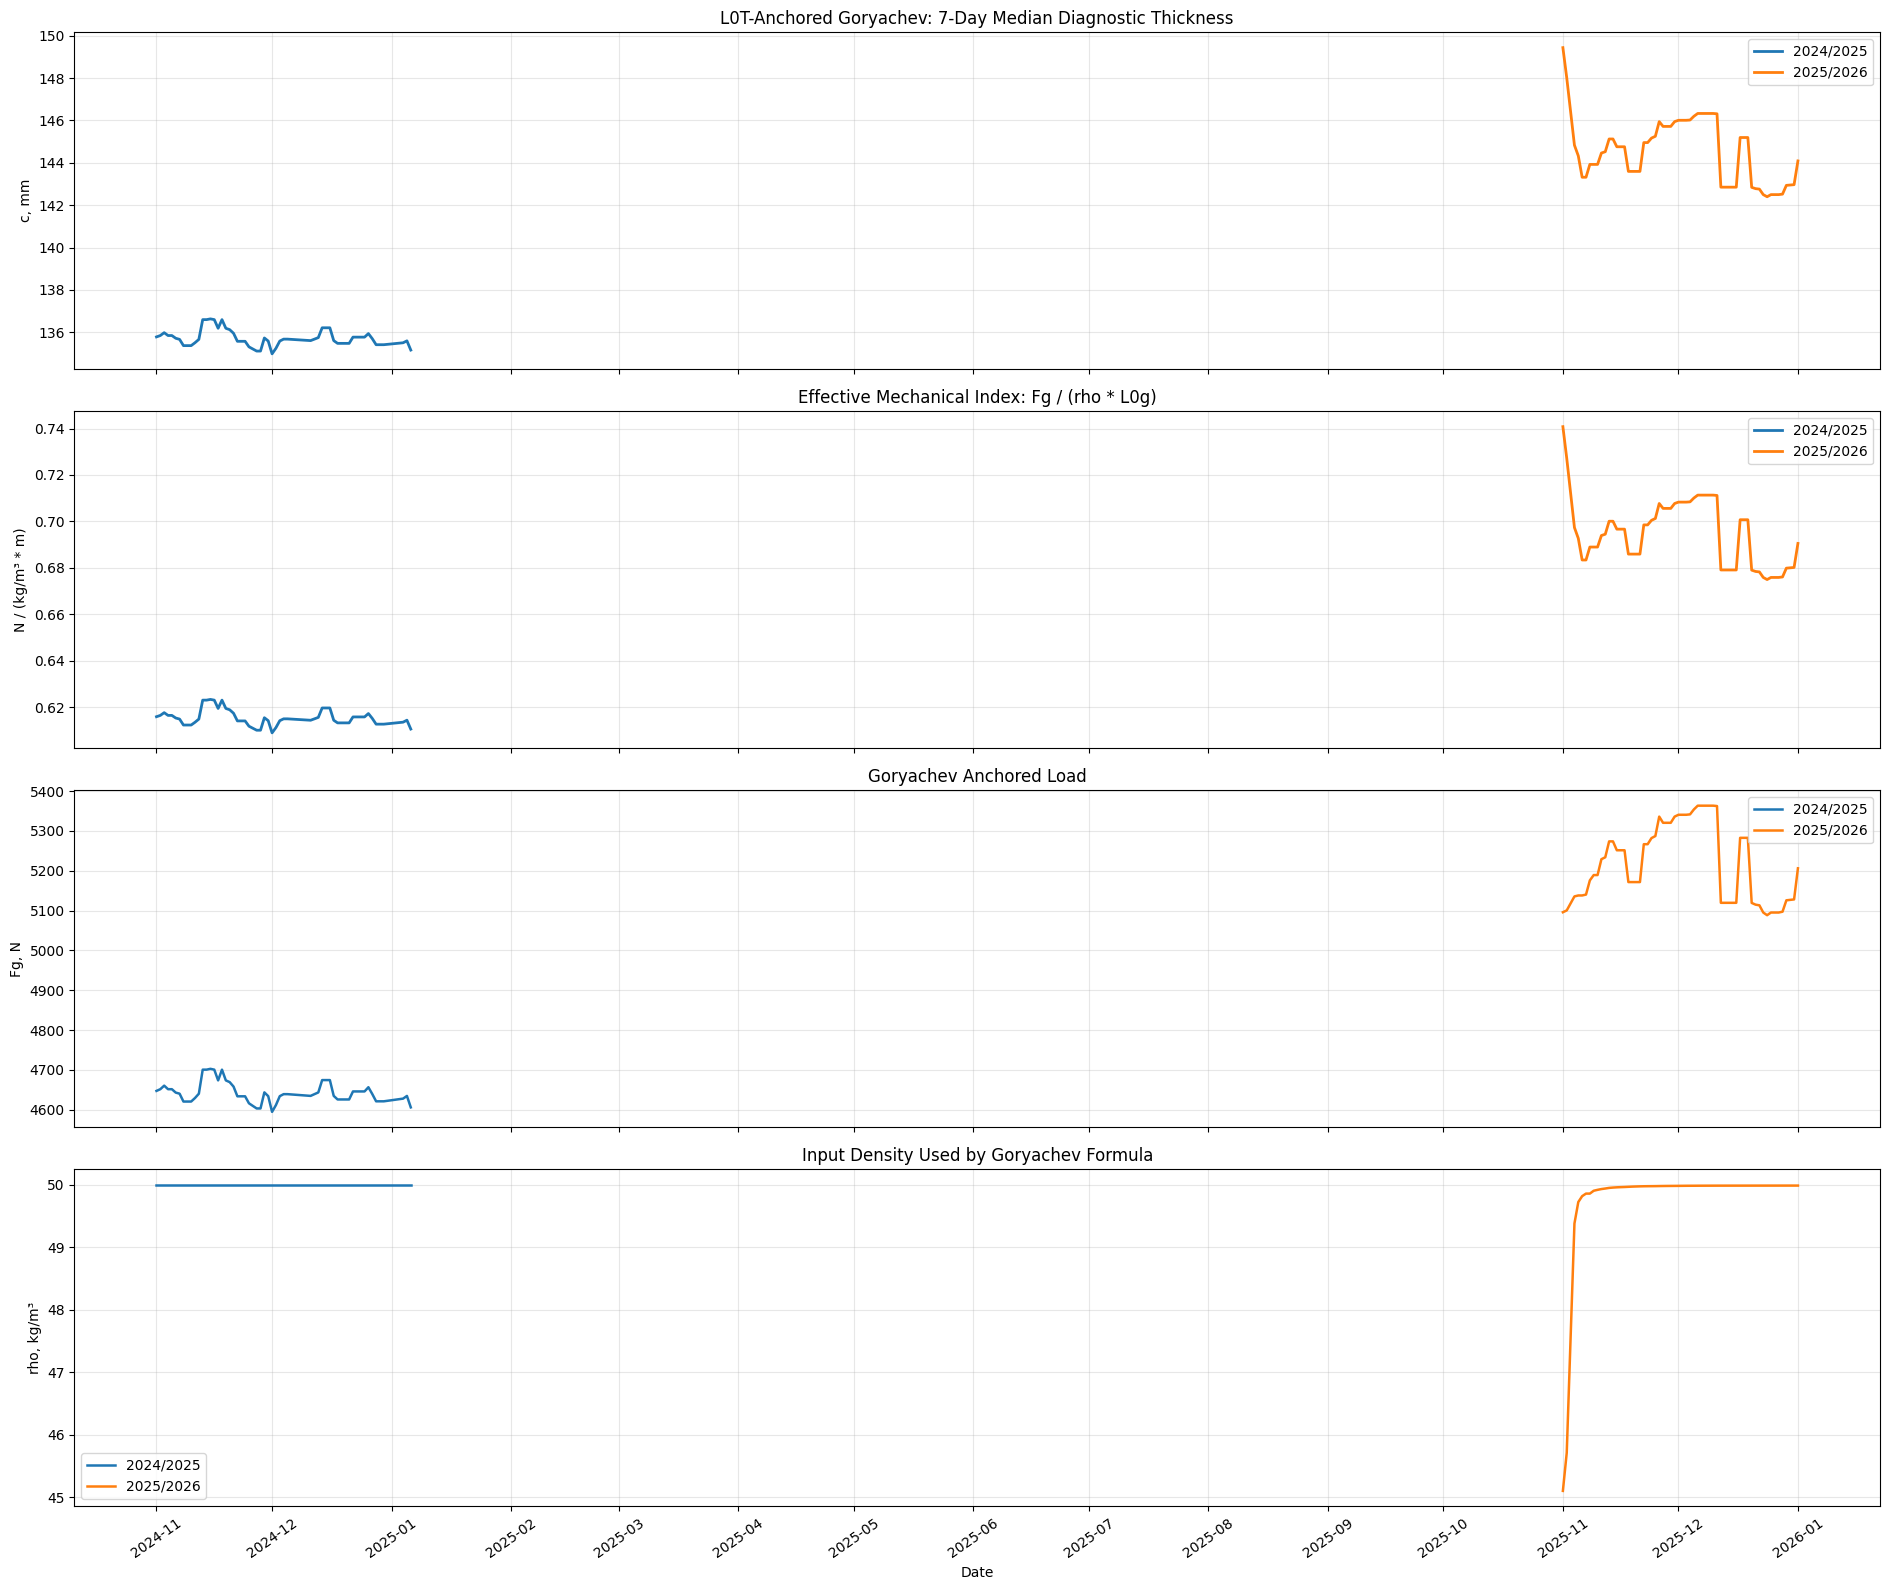

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


assert "df_gor_seasonal" in globals(), (
    "df_gor_seasonal is unavailable. "
    "Run the anchored seasonal diagnostic first."
)


required_columns = [
    "timestamp",
    "gorCmAnchoredMm",
    "gorFgAnchoredN",
    "gorL0gAnchoredM",
    "rhotkgm3",
    "phiHdeg",
    "phiK1deg",
    "isAnchoredMechanicallyValid",
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_gor_seasonal.columns
]

assert not missing_columns, (
    "Missing required columns: "
    f"{missing_columns}"
)


df_gor_drivers = (
    df_gor_seasonal
    .loc[
        df_gor_seasonal[
            "isAnchoredMechanicallyValid"
        ],
        required_columns,
    ]
    .copy()
)


df_gor_drivers["timestamp"] = pd.to_datetime(
    df_gor_drivers["timestamp"],
    errors="coerce",
)

df_gor_drivers = (
    df_gor_drivers
    .dropna(
        subset=[
            "timestamp",
            "gorCmAnchoredMm",
            "gorFgAnchoredN",
            "gorL0gAnchoredM",
            "rhotkgm3",
        ]
    )
    .sort_values(
        "timestamp"
    )
    .reset_index(
        drop=True
    )
)


df_gor_drivers["month"] = (
    df_gor_drivers["timestamp"]
    .dt.month
)

df_gor_drivers["date"] = (
    df_gor_drivers["timestamp"]
    .dt.floor(
        "D"
    )
)

df_gor_drivers["isWinter"] = (
    df_gor_drivers["month"]
    .isin(
        [
            11,
            12,
            1,
            2,
        ]
    )
)

df_gor_drivers["iceSeasonStartYear"] = np.where(
    df_gor_drivers["month"].ge(11),
    df_gor_drivers["timestamp"].dt.year,
    df_gor_drivers["timestamp"].dt.year - 1,
)


df_gor_drivers["gorMechanicalIndex"] = (
    df_gor_drivers[
        "gorFgAnchoredN"
    ]
    / (
        df_gor_drivers[
            "rhotkgm3"
        ]
        * df_gor_drivers[
            "gorL0gAnchoredM"
        ]
    )
)


df_gor_winter_drivers = (
    df_gor_drivers
    .loc[
        df_gor_drivers[
            "isWinter"
        ]
    ]
    .copy()
)


daily_goryachev_drivers = (
    df_gor_winter_drivers
    .groupby(
        [
            "iceSeasonStartYear",
            "date",
        ],
        as_index=False,
    )
    .agg(
        validRows=(
            "gorCmAnchoredMm",
            "size",
        ),
        gorCmAnchoredMm=(
            "gorCmAnchoredMm",
            "median",
        ),
        gorFgAnchoredN=(
            "gorFgAnchoredN",
            "median",
        ),
        gorL0gAnchoredM=(
            "gorL0gAnchoredM",
            "median",
        ),
        rhotkgm3=(
            "rhotkgm3",
            "median",
        ),
        phiHdeg=(
            "phiHdeg",
            "median",
        ),
        phiK1deg=(
            "phiK1deg",
            "median",
        ),
        gorMechanicalIndex=(
            "gorMechanicalIndex",
            "median",
        ),
    )
    .sort_values(
        [
            "iceSeasonStartYear",
            "date",
        ]
    )
    .reset_index(
        drop=True
    )
)


daily_goryachev_drivers[
    "seasonDay"
] = (
    daily_goryachev_drivers["date"]
    - pd.to_datetime(
        daily_goryachev_drivers[
            "iceSeasonStartYear"
        ]
        .astype(str)
        + "-11-01"
    )
).dt.days + 1


driver_columns = [
    "gorCmAnchoredMm",
    "gorFgAnchoredN",
    "gorL0gAnchoredM",
    "rhotkgm3",
    "phiHdeg",
    "phiK1deg",
    "gorMechanicalIndex",
]

for column in driver_columns:
    daily_goryachev_drivers[
        f"{column}Rolling7D"
    ] = (
        daily_goryachev_drivers
        .groupby(
            "iceSeasonStartYear"
        )[
            column
        ]
        .transform(
            lambda series: (
                series
                .rolling(
                    window=7,
                    min_periods=3,
                    center=True,
                )
                .median()
            )
        )
    )


trend_rows = []

for ice_season_year, group in daily_goryachev_drivers.groupby(
    "iceSeasonStartYear"
):
    for column in driver_columns:
        trend_group = (
            group
            .dropna(
                subset=[
                    "seasonDay",
                    column,
                ]
            )
            .copy()
        )

        if len(trend_group) < 7:
            trend_rows.append(
                {
                    "iceSeason": (
                        f"{ice_season_year}/"
                        f"{ice_season_year + 1}"
                    ),
                    "variable": column,
                    "dailyPoints": len(
                        trend_group
                    ),
                    "firstDailyMedian": np.nan,
                    "lastDailyMedian": np.nan,
                    "netChange": np.nan,
                    "trendPerDay": np.nan,
                    "trendPer30Days": np.nan,
                    "coefficientVariationPercent": np.nan,
                }
            )

            continue

        slope_per_day, intercept = np.polyfit(
            trend_group["seasonDay"],
            trend_group[column],
            deg=1,
        )

        mean_value = trend_group[
            column
        ].mean()

        std_value = trend_group[
            column
        ].std()

        trend_rows.append(
            {
                "iceSeason": (
                    f"{ice_season_year}/"
                    f"{ice_season_year + 1}"
                ),
                "variable": column,
                "dailyPoints": len(
                    trend_group
                ),
                "firstDailyMedian": (
                    trend_group[
                        column
                    ]
                    .iloc[0]
                ),
                "lastDailyMedian": (
                    trend_group[
                        column
                    ]
                    .iloc[-1]
                ),
                "netChange": (
                    trend_group[
                        column
                    ]
                    .iloc[-1]
                    - trend_group[
                        column
                    ]
                    .iloc[0]
                ),
                "trendPerDay": slope_per_day,
                "trendPer30Days": (
                    30.0
                    * slope_per_day
                ),
                "coefficientVariationPercent": (
                    100.0
                    * std_value
                    / abs(mean_value)
                    if mean_value != 0.0
                    else np.nan
                ),
            }
        )


df_gor_driver_trends = pd.DataFrame(
    trend_rows
)


correlation_rows = []

for ice_season_year, group in daily_goryachev_drivers.groupby(
    "iceSeasonStartYear"
):
    correlation_matrix = (
        group[
            driver_columns
        ]
        .corr(
            method="spearman"
        )
    )

    for variable in [
        "gorFgAnchoredN",
        "gorL0gAnchoredM",
        "rhotkgm3",
        "phiHdeg",
        "phiK1deg",
        "gorMechanicalIndex",
    ]:
        correlation_rows.append(
            {
                "iceSeason": (
                    f"{ice_season_year}/"
                    f"{ice_season_year + 1}"
                ),
                "response": "gorCmAnchoredMm",
                "predictor": variable,
                "spearmanCorrelation": (
                    correlation_matrix.loc[
                        "gorCmAnchoredMm",
                        variable,
                    ]
                ),
            }
        )


df_gor_driver_correlations = pd.DataFrame(
    correlation_rows
)


monthly_goryachev_drivers = (
    df_gor_winter_drivers
    .assign(
        monthStart=lambda frame: (
            frame["timestamp"]
            .dt.to_period("M")
            .dt.to_timestamp()
        )
    )
    .groupby(
        [
            "iceSeasonStartYear",
            "monthStart",
        ],
        as_index=False,
    )
    .agg(
        validRows=(
            "gorCmAnchoredMm",
            "size",
        ),
        gorCmAnchoredMm=(
            "gorCmAnchoredMm",
            "median",
        ),
        gorFgAnchoredN=(
            "gorFgAnchoredN",
            "median",
        ),
        gorL0gAnchoredM=(
            "gorL0gAnchoredM",
            "median",
        ),
        rhotkgm3=(
            "rhotkgm3",
            "median",
        ),
        phiHdeg=(
            "phiHdeg",
            "median",
        ),
        phiK1deg=(
            "phiK1deg",
            "median",
        ),
        gorMechanicalIndex=(
            "gorMechanicalIndex",
            "median",
        ),
    )
)


print("GORYACHEV WINTER DRIVER TRENDS")
print("=" * 100)

display(
    df_gor_driver_trends
    .sort_values(
        [
            "iceSeason",
            "variable",
        ]
    )
    .reset_index(
        drop=True
    )
)


print("\nGORYACHEV THICKNESS-DRIVER SPEARMAN CORRELATIONS")
print("=" * 100)

display(
    df_gor_driver_correlations
    .sort_values(
        [
            "iceSeason",
            "spearmanCorrelation",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)


print("\nMONTHLY GORYACHEV DRIVER MEDIANS")
print("=" * 100)

display(
    monthly_goryachev_drivers
    .sort_values(
        [
            "iceSeasonStartYear",
            "monthStart",
        ]
    )
    .reset_index(
        drop=True
    )
)


fig, axes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(19, 16),
    sharex=True,
)


for ice_season_year, group in daily_goryachev_drivers.groupby(
    "iceSeasonStartYear"
):
    label_suffix = (
        f"{ice_season_year}/"
        f"{ice_season_year + 1}"
    )

    axes[0].plot(
        group["date"],
        group[
            "gorCmAnchoredMmRolling7D"
        ],
        linewidth=2.0,
        label=label_suffix,
    )

    axes[1].plot(
        group["date"],
        group[
            "gorMechanicalIndexRolling7D"
        ],
        linewidth=2.0,
        label=label_suffix,
    )

    axes[2].plot(
        group["date"],
        group[
            "gorFgAnchoredNRolling7D"
        ],
        linewidth=1.8,
        label=label_suffix,
    )

    axes[3].plot(
        group["date"],
        group[
            "rhotkgm3Rolling7D"
        ],
        linewidth=1.8,
        label=label_suffix,
    )


axes[0].set_title(
    "L0T-Anchored Goryachev: 7-Day Median Diagnostic Thickness"
)

axes[0].set_ylabel(
    "c, mm"
)

axes[1].set_title(
    "Effective Mechanical Index: Fg / (rho * L0g)"
)

axes[1].set_ylabel(
    "N / (kg/m³ * m)"
)

axes[2].set_title(
    "Goryachev Anchored Load"
)

axes[2].set_ylabel(
    "Fg, N"
)

axes[3].set_title(
    "Input Density Used by Goryachev Formula"
)

axes[3].set_ylabel(
    "rho, kg/m³"
)

axes[3].set_xlabel(
    "Date"
)


for axis in axes:
    axis.grid(
        True,
        alpha=0.30,
    )

    axis.legend(
        loc="best"
    )


axes[3].xaxis.set_major_locator(
    mdates.MonthLocator(
        interval=1
    )
)

axes[3].xaxis.set_major_formatter(
    mdates.DateFormatter(
        "%Y-%m"
    )
)

plt.xticks(
    rotation=35
)

plt.tight_layout()
plt.show()

GORYACHEV MONTHLY COUNTERFACTUAL DECOMPOSITION


,iceSeason,monthStart,validRows,observedMonthlyMedianCmMm,formulaAtMonthlyMedianInputsMm,baselineCmMm,FgOnlyCmMm,rhoOnlyCmMm,L0gOnlyCmMm,allDriversCmMm,FgContributionMm,rhoContributionMm,L0gContributionMm,allDriversChangeMm
0,2024/2025,2024-11-01,235,135.653500,135.649942,135.649942,135.649942,135.649942,135.649942,135.649942,0.000000,0.000000e+00,0.000000,0.000000
1,2024/2025,2024-12-01,155,135.725958,135.733420,135.649942,135.719446,135.649942,135.663909,135.733420,0.069504,-1.587914e-07,0.013967,0.083478
2,2024/2025,2025-01-01,14,127.019735,127.179605,135.649942,127.161063,135.649942,135.669673,127.179605,-8.488880,-5.843049e-09,0.019731,-8.470338
3,2025/2026,2025-11-01,4198,144.672666,144.248277,144.248277,144.248277,144.248277,144.248277,144.248277,0.000000,0.000000e+00,0.000000,0.000000
4,2025/2026,2025-12-01,3458,145.195593,145.196823,144.248277,145.205221,144.217201,144.271012,145.196823,0.956944,-3.107574e-02,0.022736,0.948546
5,2025/2026,2026-01-01,17,148.159462,148.159462,144.248277,148.177744,144.215790,144.262953,148.159462,3.929467,-3.248664e-02,0.014676,3.911185


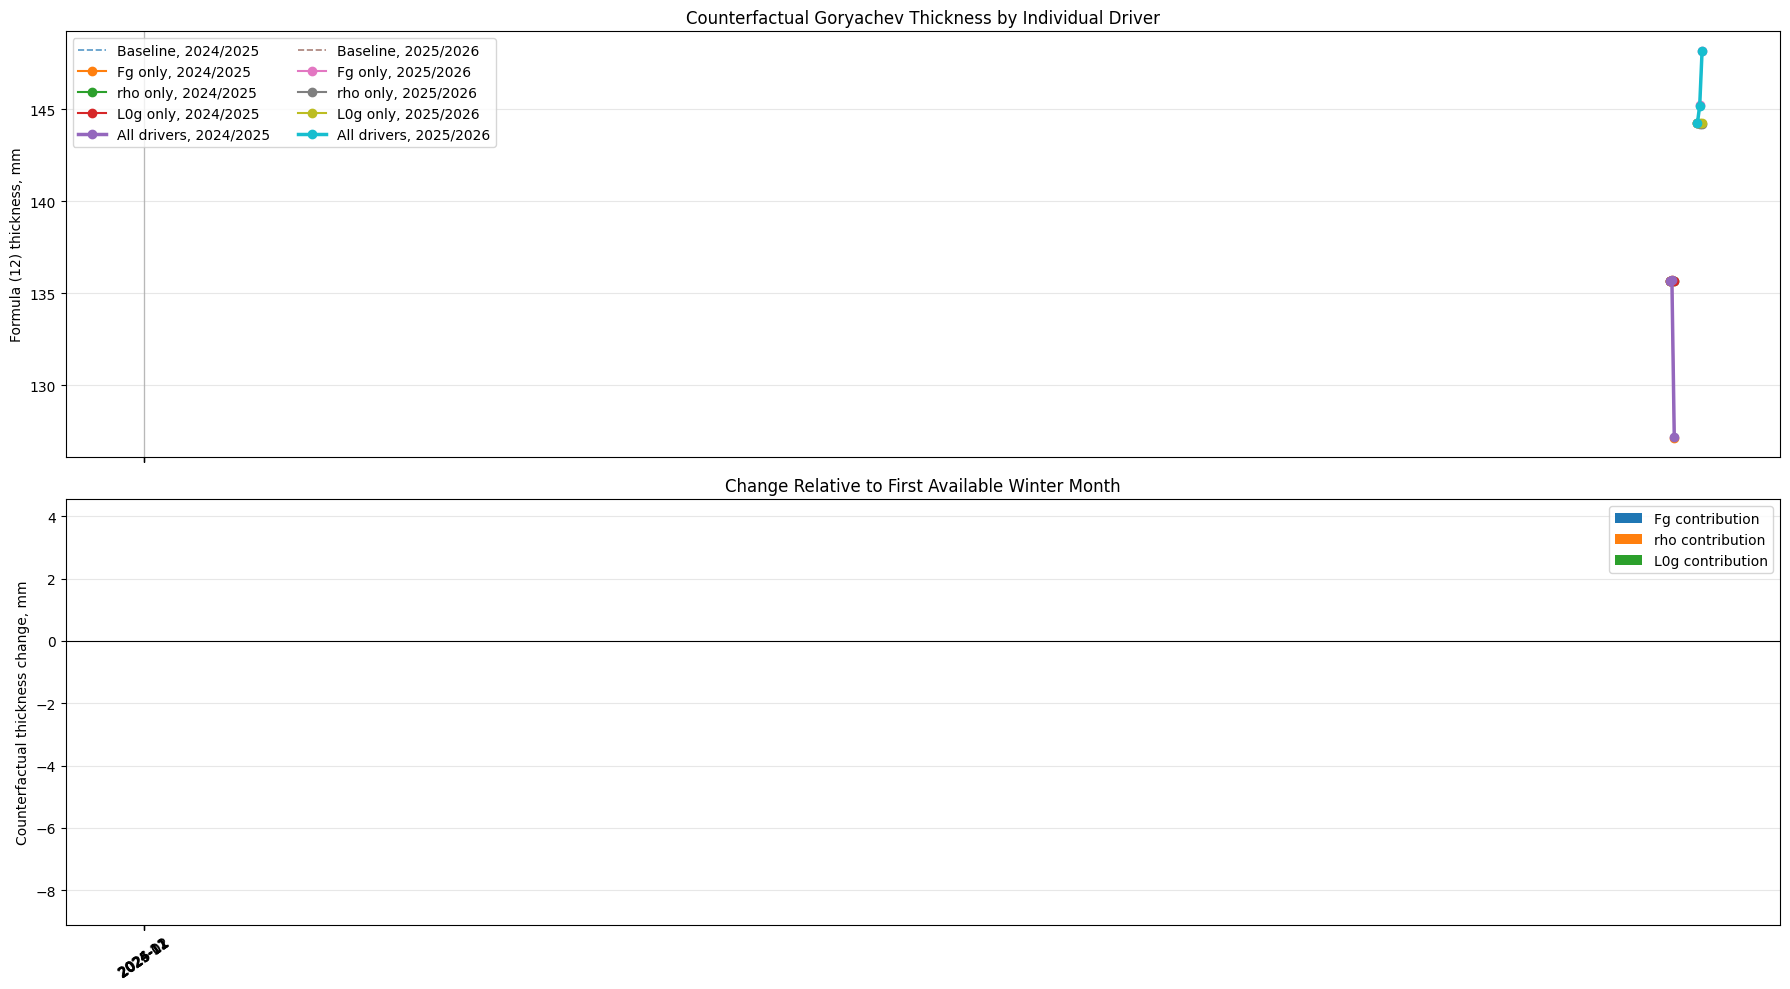

In [ ]:
from src.goryachev_model import (
    eq12_ice_wall_thickness,
)


assert "monthly_goryachev_drivers" in globals(), (
    "monthly_goryachev_drivers is unavailable. "
    "Run the Goryachev driver diagnostic first."
)

assert "cable_params" in globals(), (
    "cable_params is unavailable."
)


def resolve_dpr_m(
    parameter_object,
) -> float:
    for attribute_name in [
        "dprm",
        "dPrM",
        "D_PR_M",
    ]:
        if hasattr(
            parameter_object,
            attribute_name,
        ):
            return float(
                getattr(
                    parameter_object,
                    attribute_name,
                )
            )

    raise AttributeError(
        "Cannot resolve bare conductor diameter "
        "from cable_params."
    )


D_PR_M = resolve_dpr_m(
    cable_params
)


df_gor_counterfactual = (
    monthly_goryachev_drivers
    .copy()
    .sort_values(
        [
            "iceSeasonStartYear",
            "monthStart",
        ]
    )
    .reset_index(
        drop=True
    )
)


counterfactual_rows = []

for ice_season_year, group in df_gor_counterfactual.groupby(
    "iceSeasonStartYear"
):
    group = (
        group
        .sort_values(
            "monthStart"
        )
        .reset_index(
            drop=True
        )
    )

    if len(group) == 0:
        continue

    baseline = group.iloc[0]

    baseline_fg = float(
        baseline["gorFgAnchoredN"]
    )

    baseline_rho = float(
        baseline["rhotkgm3"]
    )

    baseline_l0g = float(
        baseline["gorL0gAnchoredM"]
    )

    baseline_cm = eq12_ice_wall_thickness(
        d_pr=D_PR_M,
        Fg=baseline_fg,
        q0g=baseline_rho,
        L0g=baseline_l0g,
    ) * 1000.0

    for _, row in group.iterrows():
        actual_fg = float(
            row["gorFgAnchoredN"]
        )

        actual_rho = float(
            row["rhotkgm3"]
        )

        actual_l0g = float(
            row["gorL0gAnchoredM"]
        )

        cm_fg_only = eq12_ice_wall_thickness(
            d_pr=D_PR_M,
            Fg=actual_fg,
            q0g=baseline_rho,
            L0g=baseline_l0g,
        ) * 1000.0

        cm_rho_only = eq12_ice_wall_thickness(
            d_pr=D_PR_M,
            Fg=baseline_fg,
            q0g=actual_rho,
            L0g=baseline_l0g,
        ) * 1000.0

        cm_l0g_only = eq12_ice_wall_thickness(
            d_pr=D_PR_M,
            Fg=baseline_fg,
            q0g=baseline_rho,
            L0g=actual_l0g,
        ) * 1000.0

        cm_all_drivers = eq12_ice_wall_thickness(
            d_pr=D_PR_M,
            Fg=actual_fg,
            q0g=actual_rho,
            L0g=actual_l0g,
        ) * 1000.0

        counterfactual_rows.append(
            {
                "iceSeason": (
                    f"{ice_season_year}/"
                    f"{ice_season_year + 1}"
                ),
                "monthStart": row[
                    "monthStart"
                ],
                "validRows": row[
                    "validRows"
                ],
                "observedMonthlyMedianCmMm": row[
                    "gorCmAnchoredMm"
                ],
                "formulaAtMonthlyMedianInputsMm": (
                    cm_all_drivers
                ),
                "baselineCmMm": baseline_cm,
                "FgOnlyCmMm": cm_fg_only,
                "rhoOnlyCmMm": cm_rho_only,
                "L0gOnlyCmMm": cm_l0g_only,
                "allDriversCmMm": cm_all_drivers,
                "FgContributionMm": (
                    cm_fg_only
                    - baseline_cm
                ),
                "rhoContributionMm": (
                    cm_rho_only
                    - baseline_cm
                ),
                "L0gContributionMm": (
                    cm_l0g_only
                    - baseline_cm
                ),
                "allDriversChangeMm": (
                    cm_all_drivers
                    - baseline_cm
                ),
            }
        )


df_gor_counterfactual = pd.DataFrame(
    counterfactual_rows
)


print("GORYACHEV MONTHLY COUNTERFACTUAL DECOMPOSITION")
print("=" * 100)

display(
    df_gor_counterfactual
    .sort_values(
        [
            "iceSeason",
            "monthStart",
        ]
    )
    .reset_index(
        drop=True
    )
)


fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(18, 10),
    sharex=True,
)


for ice_season, group in df_gor_counterfactual.groupby(
    "iceSeason"
):
    axes[0].plot(
        group["monthStart"],
        group["baselineCmMm"],
        linestyle="--",
        linewidth=1.2,
        alpha=0.75,
        label=(
            f"Baseline, {ice_season}"
        ),
    )

    axes[0].plot(
        group["monthStart"],
        group["FgOnlyCmMm"],
        marker="o",
        linewidth=1.5,
        label=(
            f"Fg only, {ice_season}"
        ),
    )

    axes[0].plot(
        group["monthStart"],
        group["rhoOnlyCmMm"],
        marker="o",
        linewidth=1.5,
        label=(
            f"rho only, {ice_season}"
        ),
    )

    axes[0].plot(
        group["monthStart"],
        group["L0gOnlyCmMm"],
        marker="o",
        linewidth=1.5,
        label=(
            f"L0g only, {ice_season}"
        ),
    )

    axes[0].plot(
        group["monthStart"],
        group["allDriversCmMm"],
        marker="o",
        linewidth=2.5,
        label=(
            f"All drivers, {ice_season}"
        ),
    )


axes[0].set_title(
    "Counterfactual Goryachev Thickness by Individual Driver"
)

axes[0].set_ylabel(
    "Formula (12) thickness, mm"
)

axes[0].grid(
    True,
    alpha=0.30,
)

axes[0].legend(
    loc="best",
    ncol=2,
)


contribution_plot = (
    df_gor_counterfactual
    .copy()
    .sort_values(
        [
            "iceSeason",
            "monthStart",
        ]
    )
)

bar_positions = np.arange(
    len(contribution_plot)
)

bar_width = 0.25

axes[1].bar(
    bar_positions - bar_width,
    contribution_plot[
        "FgContributionMm"
    ],
    width=bar_width,
    label="Fg contribution",
)

axes[1].bar(
    bar_positions,
    contribution_plot[
        "rhoContributionMm"
    ],
    width=bar_width,
    label="rho contribution",
)

axes[1].bar(
    bar_positions + bar_width,
    contribution_plot[
        "L0gContributionMm"
    ],
    width=bar_width,
    label="L0g contribution",
)

axes[1].axhline(
    0.0,
    color="black",
    linewidth=0.8,
)

axes[1].set_title(
    "Change Relative to First Available Winter Month"
)

axes[1].set_ylabel(
    "Counterfactual thickness change, mm"
)

axes[1].set_xticks(
    bar_positions
)

axes[1].set_xticklabels(
    contribution_plot[
        "monthStart"
    ]
    .dt.strftime(
        "%Y-%m"
    ),
    rotation=35,
)

axes[1].grid(
    True,
    axis="y",
    alpha=0.30,
)

axes[1].legend(
    loc="best"
)


plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


assert "df_gor_seasonal" in globals(), (
    "df_gor_seasonal is unavailable. "
    "Run the L0T-anchored seasonal diagnostic first."
)


required_columns = [
    "timestamp",
    "referenceKey",
    "gorCmAnchoredMm",
    "gorFgAnchoredN",
    "gorL0gAnchoredM",
    "phiHdeg",
    "phiK1deg",
    "referencePhiK0Deg",
    "isAnchoredMechanicallyValid",
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_gor_seasonal.columns
]

assert not missing_columns, (
    "Missing required columns: "
    f"{missing_columns}"
)


df_gor_mechanical_signal = (
    df_gor_seasonal
    .loc[
        df_gor_seasonal[
            "isAnchoredMechanicallyValid"
        ],
        required_columns,
    ]
    .copy()
)


df_gor_mechanical_signal["timestamp"] = pd.to_datetime(
    df_gor_mechanical_signal["timestamp"],
    errors="coerce",
)

df_gor_mechanical_signal = (
    df_gor_mechanical_signal
    .dropna(
        subset=[
            "timestamp",
            "referenceKey",
            "gorCmAnchoredMm",
            "gorFgAnchoredN",
            "phiHdeg",
            "phiK1deg",
            "referencePhiK0Deg",
        ]
    )
    .sort_values(
        "timestamp"
    )
    .reset_index(
        drop=True
    )
)


df_gor_mechanical_signal["month"] = (
    df_gor_mechanical_signal[
        "timestamp"
    ]
    .dt.month
)

df_gor_mechanical_signal["date"] = (
    df_gor_mechanical_signal[
        "timestamp"
    ]
    .dt.floor(
        "D"
    )
)

df_gor_mechanical_signal["weekStart"] = (
    df_gor_mechanical_signal[
        "timestamp"
    ]
    .dt.floor(
        "D"
    )
    - pd.to_timedelta(
        df_gor_mechanical_signal[
            "timestamp"
        ]
        .dt.weekday,
        unit="D",
    )
)

df_gor_mechanical_signal["isWinter"] = (
    df_gor_mechanical_signal[
        "month"
    ]
    .isin(
        [
            11,
            12,
            1,
            2,
        ]
    )
)

df_gor_mechanical_signal["iceSeasonStartYear"] = np.where(
    df_gor_mechanical_signal[
        "month"
    ]
    .ge(11),
    df_gor_mechanical_signal[
        "timestamp"
    ]
    .dt.year,
    df_gor_mechanical_signal[
        "timestamp"
    ]
    .dt.year - 1,
)


df_gor_mechanical_signal[
    "deltaPhiKDeg"
] = (
    df_gor_mechanical_signal[
        "phiK1deg"
    ]
    - df_gor_mechanical_signal[
        "referencePhiK0Deg"
    ]
)


df_gor_winter_mechanical = (
    df_gor_mechanical_signal
    .loc[
        df_gor_mechanical_signal[
            "isWinter"
        ]
    ]
    .copy()
)


df_gor_winter_mechanical[
    "seasonDay"
] = (
    df_gor_winter_mechanical[
        "date"
    ]
    - pd.to_datetime(
        df_gor_winter_mechanical[
            "iceSeasonStartYear"
        ]
        .astype(str)
        + "-11-01"
    )
).dt.days + 1


df_gor_winter_mechanical[
    "winterPhase"
] = np.select(
    [
        df_gor_winter_mechanical[
            "seasonDay"
        ]
        .between(
            1,
            30,
        ),
        df_gor_winter_mechanical[
            "seasonDay"
        ]
        .between(
            31,
            61,
        ),
        df_gor_winter_mechanical[
            "seasonDay"
        ]
        .ge(62),
    ],
    [
        "early_days_1_30_Nov",
        "middle_days_31_61_Dec",
        "late_days_62_123_Jan_Feb",
    ],
    default="outside_expected_window",
)


daily_mechanical_signal = (
    df_gor_winter_mechanical
    .groupby(
        [
            "iceSeasonStartYear",
            "date",
        ],
        as_index=False,
    )
    .agg(
        validRows=(
            "gorCmAnchoredMm",
            "size",
        ),
        referenceKeyNunique=(
            "referenceKey",
            "nunique",
        ),
        referenceKey=(
            "referenceKey",
            "first",
        ),
        phiHdeg=(
            "phiHdeg",
            "median",
        ),
        phiK1deg=(
            "phiK1deg",
            "median",
        ),
        referencePhiK0Deg=(
            "referencePhiK0Deg",
            "median",
        ),
        deltaPhiKDeg=(
            "deltaPhiKDeg",
            "median",
        ),
        gorFgAnchoredN=(
            "gorFgAnchoredN",
            "median",
        ),
        gorCmAnchoredMm=(
            "gorCmAnchoredMm",
            "median",
        ),
        gorL0gAnchoredM=(
            "gorL0gAnchoredM",
            "median",
        ),
    )
    .sort_values(
        [
            "iceSeasonStartYear",
            "date",
        ]
    )
    .reset_index(
        drop=True
    )
)


daily_mechanical_signal[
    "seasonDay"
] = (
    daily_mechanical_signal[
        "date"
    ]
    - pd.to_datetime(
        daily_mechanical_signal[
            "iceSeasonStartYear"
        ]
        .astype(str)
        + "-11-01"
    )
).dt.days + 1


daily_mechanical_signal[
    "winterPhase"
] = np.select(
    [
        daily_mechanical_signal[
            "seasonDay"
        ]
        .between(
            1,
            30,
        ),
        daily_mechanical_signal[
            "seasonDay"
        ]
        .between(
            31,
            61,
        ),
        daily_mechanical_signal[
            "seasonDay"
        ]
        .ge(62),
    ],
    [
        "early_days_1_30_Nov",
        "middle_days_31_61_Dec",
        "late_days_62_123_Jan_Feb",
    ],
    default="outside_expected_window",
)


rolling_columns = [
    "phiHdeg",
    "phiK1deg",
    "deltaPhiKDeg",
    "gorFgAnchoredN",
    "gorCmAnchoredMm",
]

for column in rolling_columns:
    daily_mechanical_signal[
        f"{column}Rolling7D"
    ] = (
        daily_mechanical_signal
        .groupby(
            "iceSeasonStartYear"
        )[
            column
        ]
        .transform(
            lambda series: (
                series
                .rolling(
                    window=7,
                    min_periods=3,
                    center=True,
                )
                .median()
            )
        )
    )


weekly_mechanical_signal = (
    df_gor_winter_mechanical
    .groupby(
        [
            "iceSeasonStartYear",
            "weekStart",
        ],
        as_index=False,
    )
    .agg(
        validRows=(
            "gorCmAnchoredMm",
            "size",
        ),
        referenceKeyNunique=(
            "referenceKey",
            "nunique",
        ),
        phiHdeg=(
            "phiHdeg",
            "median",
        ),
        phiK1deg=(
            "phiK1deg",
            "median",
        ),
        referencePhiK0Deg=(
            "referencePhiK0Deg",
            "median",
        ),
        deltaPhiKDeg=(
            "deltaPhiKDeg",
            "median",
        ),
        gorFgAnchoredN=(
            "gorFgAnchoredN",
            "median",
        ),
        gorCmAnchoredMm=(
            "gorCmAnchoredMm",
            "median",
        ),
    )
    .sort_values(
        [
            "iceSeasonStartYear",
            "weekStart",
        ]
    )
    .reset_index(
        drop=True
    )
)


phase_mechanical_summary = (
    df_gor_winter_mechanical
    .groupby(
        [
            "iceSeasonStartYear",
            "winterPhase",
        ],
        as_index=False,
    )
    .agg(
        validRows=(
            "gorCmAnchoredMm",
            "size",
        ),
        activeDays=(
            "date",
            "nunique",
        ),
        referenceKeyNunique=(
            "referenceKey",
            "nunique",
        ),
        phiHdegMedian=(
            "phiHdeg",
            "median",
        ),
        phiK1degMedian=(
            "phiK1deg",
            "median",
        ),
        phiK1degP05=(
            "phiK1deg",
            lambda series: series.quantile(
                0.05
            ),
        ),
        phiK1degP95=(
            "phiK1deg",
            lambda series: series.quantile(
                0.95
            ),
        ),
        deltaPhiKDegMedian=(
            "deltaPhiKDeg",
            "median",
        ),
        deltaPhiKDegP05=(
            "deltaPhiKDeg",
            lambda series: series.quantile(
                0.05
            ),
        ),
        deltaPhiKDegP95=(
            "deltaPhiKDeg",
            lambda series: series.quantile(
                0.95
            ),
        ),
        gorFgMedianN=(
            "gorFgAnchoredN",
            "median",
        ),
        gorFgP05N=(
            "gorFgAnchoredN",
            lambda series: series.quantile(
                0.05
            ),
        ),
        gorFgP95N=(
            "gorFgAnchoredN",
            lambda series: series.quantile(
                0.95
            ),
        ),
        gorCmMedianMm=(
            "gorCmAnchoredMm",
            "median",
        ),
        gorCmP05Mm=(
            "gorCmAnchoredMm",
            lambda series: series.quantile(
                0.05
            ),
        ),
        gorCmP95Mm=(
            "gorCmAnchoredMm",
            lambda series: series.quantile(
                0.95
            ),
        ),
    )
    .sort_values(
        [
            "iceSeasonStartYear",
            "winterPhase",
        ]
    )
    .reset_index(
        drop=True
    )
)


reference_key_summary = (
    df_gor_winter_mechanical
    .groupby(
        [
            "iceSeasonStartYear",
            "referenceKey",
        ],
        as_index=False,
    )
    .agg(
        validRows=(
            "gorCmAnchoredMm",
            "size",
        ),
        firstTimestamp=(
            "timestamp",
            "min",
        ),
        lastTimestamp=(
            "timestamp",
            "max",
        ),
        activeDays=(
            "date",
            "nunique",
        ),
        phiK1MedianDeg=(
            "phiK1deg",
            "median",
        ),
        deltaPhiKMedianDeg=(
            "deltaPhiKDeg",
            "median",
        ),
        FgMedianN=(
            "gorFgAnchoredN",
            "median",
        ),
        CmMedianMm=(
            "gorCmAnchoredMm",
            "median",
        ),
    )
    .sort_values(
        [
            "iceSeasonStartYear",
            "firstTimestamp",
        ]
    )
    .reset_index(
        drop=True
    )
)


correlation_rows = []

for ice_season_year, group in daily_mechanical_signal.groupby(
    "iceSeasonStartYear"
):
    correlation_matrix = (
        group[
            [
                "phiHdeg",
                "phiK1deg",
                "deltaPhiKDeg",
                "gorFgAnchoredN",
                "gorCmAnchoredMm",
            ]
        ]
        .corr(
            method="spearman"
        )
    )

    for predictor in [
        "phiHdeg",
        "phiK1deg",
        "deltaPhiKDeg",
        "gorFgAnchoredN",
    ]:
        correlation_rows.append(
            {
                "iceSeason": (
                    f"{ice_season_year}/"
                    f"{ice_season_year + 1}"
                ),
                "response": "gorFgAnchoredN",
                "predictor": predictor,
                "spearmanCorrelation": (
                    correlation_matrix.loc[
                        "gorFgAnchoredN",
                        predictor,
                    ]
                ),
            }
        )

        correlation_rows.append(
            {
                "iceSeason": (
                    f"{ice_season_year}/"
                    f"{ice_season_year + 1}"
                ),
                "response": "gorCmAnchoredMm",
                "predictor": predictor,
                "spearmanCorrelation": (
                    correlation_matrix.loc[
                        "gorCmAnchoredMm",
                        predictor,
                    ]
                ),
            }
        )


df_gor_mechanical_correlations = pd.DataFrame(
    correlation_rows
)


print("GORYACHEV WINTER PHASE MECHANICAL SUMMARY")
print("=" * 100)

display(
    phase_mechanical_summary
)


print("\nGORYACHEV WINTER REFERENCE-KEY COVERAGE")
print("=" * 100)

display(
    reference_key_summary
)


print("\nGORYACHEV MECHANICAL CHAIN SPEARMAN CORRELATIONS")
print("=" * 100)

display(
    df_gor_mechanical_correlations
    .sort_values(
        [
            "iceSeason",
            "response",
            "spearmanCorrelation",
        ],
        ascending=[
            True,
            True,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)


print("\nWEEKLY ROBUST MECHANICAL SIGNAL")
print("=" * 100)

display(
    weekly_mechanical_signal
)

GORYACHEV WINTER PHASE MECHANICAL SUMMARY


,iceSeasonStartYear,winterPhase,validRows,activeDays,referenceKeyNunique,phiHdegMedian,phiK1degMedian,phiK1degP05,phiK1degP95,deltaPhiKDegMedian,deltaPhiKDegP05,deltaPhiKDegP95,gorFgMedianN,gorFgP05N,gorFgP95N,gorCmMedianMm,gorCmP05Mm,gorCmP95Mm
0,2024,early_days_1_30_Nov,235,30,1,2.555,-3.815,-4.0680,-3.5320,10.496095,10.243095,10.779095,4638.331146,4526.236738,4764.042408,135.653500,133.927208,137.564055
1,2024,late_days_62_123_Jan_Feb,14,3,1,2.435,-5.040,-7.3120,-3.4325,9.271095,6.999095,10.878595,4097.062909,3093.140356,4807.301605,127.019735,109.788882,138.215048
2,2024,middle_days_31_61_Dec,155,25,1,2.545,-3.805,-3.9815,-3.5385,10.506095,10.329595,10.772595,4642.901185,4565.094139,4761.253059,135.725958,134.546558,137.522080
3,2025,early_days_1_30_Nov,4198,30,1,2.685,-3.585,-3.9350,-3.2050,11.800714,11.450714,12.180714,5216.097528,5060.314651,5384.300633,144.672666,142.383742,150.784487
4,2025,late_days_62_123_Jan_Feb,17,1,1,1.945,-2.955,-3.4850,-2.6610,12.430714,11.900714,12.724714,5493.461070,5259.960120,5623.099474,148.159462,144.862951,149.957105
5,2025,middle_days_31_61_Dec,3458,31,1,2.640,-3.435,-4.1350,-2.7150,11.950714,11.250714,12.670714,5282.983096,4973.658763,5600.710796,145.195593,140.721409,149.666796



GORYACHEV WINTER REFERENCE-KEY COVERAGE


,iceSeasonStartYear,referenceKey,validRows,firstTimestamp,lastTimestamp,activeDays,phiK1MedianDeg,deltaPhiKMedianDeg,FgMedianN,CmMedianMm
0,2024,1|2024-10,404,2024-11-01 05:08:42,2025-01-06 04:28:33,58,-3.8125,10.498595,4640.180961,135.701363
1,2025,3|2025-10,7673,2025-11-01 00:10:28,2026-01-01 03:05:53,62,-3.5350,11.850714,5237.889810,144.802523



GORYACHEV MECHANICAL CHAIN SPEARMAN CORRELATIONS


,iceSeason,response,predictor,spearmanCorrelation
0,2024/2025,gorCmAnchoredMm,gorFgAnchoredN,0.999385
1,2024/2025,gorCmAnchoredMm,phiK1deg,0.999031
2,2024/2025,gorCmAnchoredMm,deltaPhiKDeg,0.999015
3,2024/2025,gorCmAnchoredMm,phiHdeg,0.231365
4,2024/2025,gorFgAnchoredN,gorFgAnchoredN,1.000000
5,2024/2025,gorFgAnchoredN,phiK1deg,0.999154
6,2024/2025,gorFgAnchoredN,deltaPhiKDeg,0.999108
7,2024/2025,gorFgAnchoredN,phiHdeg,0.241211
8,2025/2026,gorCmAnchoredMm,phiK1deg,0.809144
9,2025/2026,gorCmAnchoredMm,deltaPhiKDeg,0.809144



WEEKLY ROBUST MECHANICAL SIGNAL


,iceSeasonStartYear,weekStart,validRows,referenceKeyNunique,phiHdeg,phiK1deg,referencePhiK0Deg,deltaPhiKDeg,gorFgAnchoredN,gorCmAnchoredMm
0,2024,2024-10-28,22,1,2.495,-3.840,-14.311095,10.471095,4627.055155,135.474140
1,2024,2024-11-04,48,1,2.555,-3.830,-14.311095,10.481095,4631.431632,135.535967
2,2024,2024-11-11,51,1,2.520,-3.715,-14.311095,10.596095,4682.539847,136.328771
3,2024,2024-11-18,57,1,2.445,-3.785,-14.311095,10.526095,4651.685039,135.857012
4,2024,2024-11-25,65,1,2.735,-3.885,-14.311095,10.426095,4607.842055,135.186449
5,2024,2024-12-02,27,1,2.545,-3.805,-14.311095,10.506095,4642.373596,135.715765
6,2024,2024-12-09,28,1,2.580,-3.790,-14.311095,10.521095,4649.994930,135.847832
7,2024,2024-12-16,48,1,2.530,-3.815,-14.311095,10.496095,4638.792009,135.669290
8,2024,2024-12-23,42,1,2.520,-3.810,-14.311095,10.501095,4641.021772,135.704908
9,2024,2024-12-30,14,1,2.435,-5.040,-14.311095,9.271095,4097.062909,127.019735


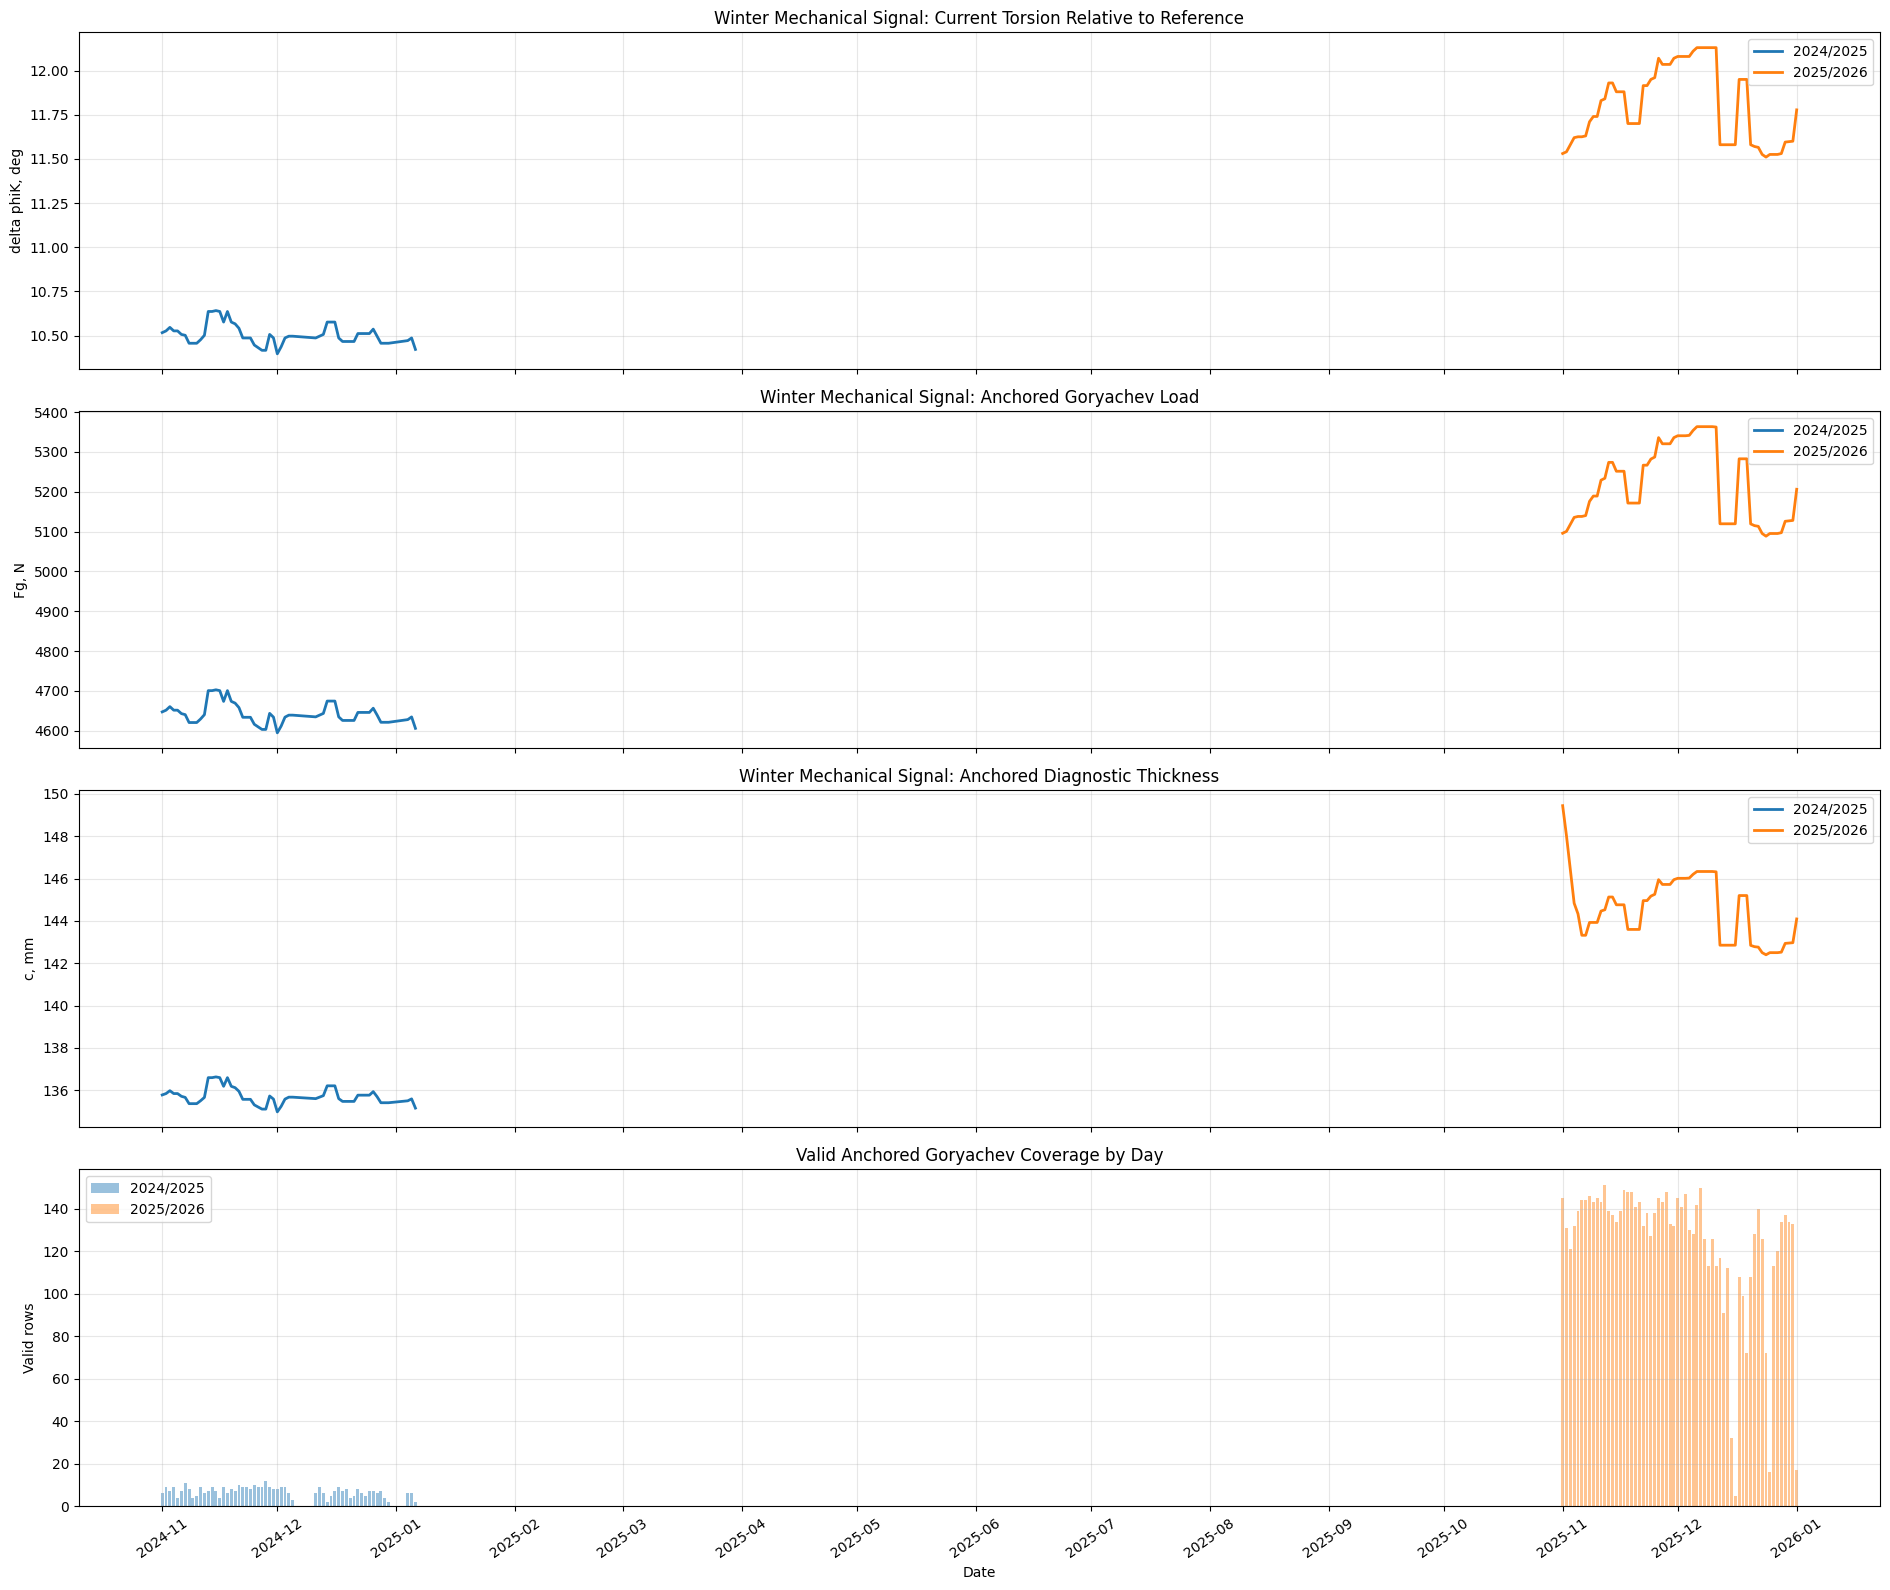

In [ ]:
fig, axes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(19, 16),
    sharex=True,
)


for ice_season_year, group in daily_mechanical_signal.groupby(
    "iceSeasonStartYear"
):
    season_label = (
        f"{ice_season_year}/"
        f"{ice_season_year + 1}"
    )

    axes[0].plot(
        group["date"],
        group[
            "deltaPhiKDegRolling7D"
        ],
        linewidth=2.0,
        label=season_label,
    )

    axes[1].plot(
        group["date"],
        group[
            "gorFgAnchoredNRolling7D"
        ],
        linewidth=2.0,
        label=season_label,
    )

    axes[2].plot(
        group["date"],
        group[
            "gorCmAnchoredMmRolling7D"
        ],
        linewidth=2.0,
        label=season_label,
    )

    axes[3].bar(
        group["date"],
        group["validRows"],
        alpha=0.45,
        width=0.75,
        label=season_label,
    )


axes[0].set_title(
    "Winter Mechanical Signal: Current Torsion Relative to Reference"
)

axes[0].set_ylabel(
    "delta phiK, deg"
)

axes[1].set_title(
    "Winter Mechanical Signal: Anchored Goryachev Load"
)

axes[1].set_ylabel(
    "Fg, N"
)

axes[2].set_title(
    "Winter Mechanical Signal: Anchored Diagnostic Thickness"
)

axes[2].set_ylabel(
    "c, mm"
)

axes[3].set_title(
    "Valid Anchored Goryachev Coverage by Day"
)

axes[3].set_ylabel(
    "Valid rows"
)

axes[3].set_xlabel(
    "Date"
)


for axis in axes:
    axis.grid(
        True,
        alpha=0.30,
    )

    axis.legend(
        loc="best"
    )


axes[3].xaxis.set_major_locator(
    mdates.MonthLocator(
        interval=1
    )
)

axes[3].xaxis.set_major_formatter(
    mdates.DateFormatter(
        "%Y-%m"
    )
)

plt.xticks(
    rotation=35
)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd


assert "df_goryachev_reference_states" in globals(), (
    "df_goryachev_reference_states is unavailable."
)

assert "df_gor_winter_mechanical" in globals(), (
    "df_gor_winter_mechanical is unavailable. "
    "Run the winter mechanical signal diagnostic first."
)


REFERENCE_KEY_COLUMN = "goryachevReferenceKey"

assert REFERENCE_KEY_COLUMN in (
    df_goryachev_reference_states.columns
), (
    "goryachevReferenceKey is absent from "
    "df_goryachev_reference_states."
)


required_reference_columns = [
    REFERENCE_KEY_COLUMN,
    "phiHcalDeg",
    "phiK1calDeg",
    "phiK0calDeg",
    "FgCalN",
]

missing_reference_columns = [
    column
    for column in required_reference_columns
    if column not in df_goryachev_reference_states.columns
]

assert not missing_reference_columns, (
    "Reference table is missing columns: "
    f"{missing_reference_columns}"
)


df_reference_geometry = (
    df_goryachev_reference_states[
        required_reference_columns
    ]
    .copy()
    .rename(
        columns={
            REFERENCE_KEY_COLUMN: "referenceKey",
            "phiHcalDeg": "referencePhiHCalDeg",
            "phiK1calDeg": "referencePhiK1CalDeg",
            "phiK0calDeg": "referencePhiK0CalDeg",
            "FgCalN": "referenceFgCalN",
        }
    )
)


df_gor_raw_sensor_reference = (
    df_gor_winter_mechanical
    .merge(
        df_reference_geometry,
        on="referenceKey",
        how="left",
        validate="many_to_one",
    )
    .copy()
)


assert (
    df_gor_raw_sensor_reference[
        "referencePhiHCalDeg"
    ]
    .notna()
    .all()
), (
    "Some winter rows failed to join "
    "the reference geometry table."
)


df_gor_raw_sensor_reference[
    "deltaPhiHSensorDeg"
] = (
    df_gor_raw_sensor_reference[
        "phiHdeg"
    ]
    - df_gor_raw_sensor_reference[
        "referencePhiHCalDeg"
    ]
)


df_gor_raw_sensor_reference[
    "deltaPhiKSensorDeg"
] = (
    df_gor_raw_sensor_reference[
        "phiK1deg"
    ]
    - df_gor_raw_sensor_reference[
        "referencePhiK1CalDeg"
    ]
)


df_gor_raw_sensor_reference[
    "derivedMinusRawKOffsetDeg"
] = (
    df_gor_raw_sensor_reference[
        "referencePhiK1CalDeg"
    ]
    - df_gor_raw_sensor_reference[
        "referencePhiK0CalDeg"
    ]
)


raw_reference_phase_summary = (
    df_gor_raw_sensor_reference
    .groupby(
        [
            "iceSeasonStartYear",
            "winterPhase",
        ],
        as_index=False,
    )
    .agg(
        validRows=(
            "gorCmAnchoredMm",
            "size",
        ),
        activeDays=(
            "date",
            "nunique",
        ),
        referenceKey=(
            "referenceKey",
            "first",
        ),
        phiHCurrentMedianDeg=(
            "phiHdeg",
            "median",
        ),
        phiHCalibrationMedianDeg=(
            "referencePhiHCalDeg",
            "median",
        ),
        deltaPhiHSensorMedianDeg=(
            "deltaPhiHSensorDeg",
            "median",
        ),
        phiK1CurrentMedianDeg=(
            "phiK1deg",
            "median",
        ),
        phiK1CalibrationMedianDeg=(
            "referencePhiK1CalDeg",
            "median",
        ),
        deltaPhiKSensorMedianDeg=(
            "deltaPhiKSensorDeg",
            "median",
        ),
        phiK0DerivedMedianDeg=(
            "referencePhiK0CalDeg",
            "median",
        ),
        deltaPhiKDerivedMedianDeg=(
            "deltaPhiKDeg",
            "median",
        ),
        derivedMinusRawKOffsetDeg=(
            "derivedMinusRawKOffsetDeg",
            "median",
        ),
        FgMedianN=(
            "gorFgAnchoredN",
            "median",
        ),
        CmMedianMm=(
            "gorCmAnchoredMm",
            "median",
        ),
    )
    .sort_values(
        [
            "iceSeasonStartYear",
            "winterPhase",
        ]
    )
    .reset_index(
        drop=True
    )
)


raw_reference_monthly_summary = (
    df_gor_raw_sensor_reference
    .assign(
        monthStart=lambda frame: (
            frame["date"]
            .dt.to_period("M")
            .dt.to_timestamp()
        )
    )
    .groupby(
        [
            "iceSeasonStartYear",
            "monthStart",
        ],
        as_index=False,
    )
    .agg(
        validRows=(
            "gorCmAnchoredMm",
            "size",
        ),
        referenceKey=(
            "referenceKey",
            "first",
        ),
        deltaPhiHSensorMedianDeg=(
            "deltaPhiHSensorDeg",
            "median",
        ),
        deltaPhiKSensorMedianDeg=(
            "deltaPhiKSensorDeg",
            "median",
        ),
        deltaPhiKDerivedMedianDeg=(
            "deltaPhiKDeg",
            "median",
        ),
        FgMedianN=(
            "gorFgAnchoredN",
            "median",
        ),
        CmMedianMm=(
            "gorCmAnchoredMm",
            "median",
        ),
    )
    .sort_values(
        [
            "iceSeasonStartYear",
            "monthStart",
        ]
    )
    .reset_index(
        drop=True
    )
)


raw_reference_correlations = []

for ice_season_year, group in df_gor_raw_sensor_reference.groupby(
    "iceSeasonStartYear"
):
    correlation_frame = group[
        [
            "deltaPhiHSensorDeg",
            "deltaPhiKSensorDeg",
            "deltaPhiKDeg",
            "gorFgAnchoredN",
            "gorCmAnchoredMm",
        ]
    ]

    correlation_matrix = correlation_frame.corr(
        method="spearman"
    )

    for predictor in [
        "deltaPhiHSensorDeg",
        "deltaPhiKSensorDeg",
        "deltaPhiKDeg",
    ]:
        raw_reference_correlations.append(
            {
                "iceSeason": (
                    f"{ice_season_year}/"
                    f"{ice_season_year + 1}"
                ),
                "response": "gorFgAnchoredN",
                "predictor": predictor,
                "spearmanCorrelation": (
                    correlation_matrix.loc[
                        "gorFgAnchoredN",
                        predictor,
                    ]
                ),
            }
        )

        raw_reference_correlations.append(
            {
                "iceSeason": (
                    f"{ice_season_year}/"
                    f"{ice_season_year + 1}"
                ),
                "response": "gorCmAnchoredMm",
                "predictor": predictor,
                "spearmanCorrelation": (
                    correlation_matrix.loc[
                        "gorCmAnchoredMm",
                        predictor,
                    ]
                ),
            }
        )


df_gor_raw_reference_correlations = pd.DataFrame(
    raw_reference_correlations
)


print("RAW SENSOR VS DERIVED REFERENCE PHASE SUMMARY")
print("=" * 100)

display(
    raw_reference_phase_summary
)


print("\nRAW SENSOR VS DERIVED REFERENCE MONTHLY SUMMARY")
print("=" * 100)

display(
    raw_reference_monthly_summary
)


print("\nRAW SENSOR VS DERIVED REFERENCE CORRELATIONS")
print("=" * 100)

display(
    df_gor_raw_reference_correlations
    .sort_values(
        [
            "iceSeason",
            "response",
            "spearmanCorrelation",
        ],
        ascending=[
            True,
            True,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)

RAW SENSOR VS DERIVED REFERENCE PHASE SUMMARY


,iceSeasonStartYear,winterPhase,validRows,activeDays,referenceKey,phiHCurrentMedianDeg,phiHCalibrationMedianDeg,deltaPhiHSensorMedianDeg,phiK1CurrentMedianDeg,phiK1CalibrationMedianDeg,deltaPhiKSensorMedianDeg,phiK0DerivedMedianDeg,deltaPhiKDerivedMedianDeg,derivedMinusRawKOffsetDeg,FgMedianN,CmMedianMm
0,2024,early_days_1_30_Nov,235,30,1|2024-10,2.555,2.525,0.030,-3.815,-3.835,0.020,-14.311095,10.496095,10.476095,4638.331146,135.653500
1,2024,late_days_62_123_Jan_Feb,14,3,1|2024-10,2.435,2.525,-0.090,-5.040,-3.835,-1.205,-14.311095,9.271095,10.476095,4097.062909,127.019735
2,2024,middle_days_31_61_Dec,155,25,1|2024-10,2.545,2.525,0.020,-3.805,-3.835,0.030,-14.311095,10.506095,10.476095,4642.901185,135.725958
3,2025,early_days_1_30_Nov,4198,30,3|2025-10,2.685,2.355,0.330,-3.585,-4.155,0.570,-15.385714,11.800714,11.230714,5216.097528,144.672666
4,2025,late_days_62_123_Jan_Feb,17,1,3|2025-10,1.945,2.355,-0.410,-2.955,-4.155,1.200,-15.385714,12.430714,11.230714,5493.461070,148.159462
5,2025,middle_days_31_61_Dec,3458,31,3|2025-10,2.640,2.355,0.285,-3.435,-4.155,0.720,-15.385714,11.950714,11.230714,5282.983096,145.195593



RAW SENSOR VS DERIVED REFERENCE MONTHLY SUMMARY


,iceSeasonStartYear,monthStart,validRows,referenceKey,deltaPhiHSensorMedianDeg,deltaPhiKSensorMedianDeg,deltaPhiKDerivedMedianDeg,FgMedianN,CmMedianMm
0,2024,2024-11-01,235,1|2024-10,0.030,0.020,10.496095,4638.331146,135.653500
1,2024,2024-12-01,155,1|2024-10,0.020,0.030,10.506095,4642.901185,135.725958
2,2024,2025-01-01,14,1|2024-10,-0.090,-1.205,9.271095,4097.062909,127.019735
3,2025,2025-11-01,4198,3|2025-10,0.330,0.570,11.800714,5216.097528,144.672666
4,2025,2025-12-01,3458,3|2025-10,0.285,0.720,11.950714,5282.983096,145.195593
5,2025,2026-01-01,17,3|2025-10,-0.410,1.200,12.430714,5493.461070,148.159462



RAW SENSOR VS DERIVED REFERENCE CORRELATIONS


,iceSeason,response,predictor,spearmanCorrelation
0,2024/2025,gorCmAnchoredMm,deltaPhiKDeg,0.999672
1,2024/2025,gorCmAnchoredMm,deltaPhiKSensorDeg,0.999581
2,2024/2025,gorCmAnchoredMm,deltaPhiHSensorDeg,0.132370
3,2024/2025,gorFgAnchoredN,deltaPhiKDeg,0.999688
4,2024/2025,gorFgAnchoredN,deltaPhiKSensorDeg,0.999618
5,2024/2025,gorFgAnchoredN,deltaPhiHSensorDeg,0.138148
6,2025/2026,gorCmAnchoredMm,deltaPhiKDeg,0.830091
7,2025/2026,gorCmAnchoredMm,deltaPhiKSensorDeg,0.829988
8,2025/2026,gorCmAnchoredMm,deltaPhiHSensorDeg,0.342393
9,2025/2026,gorFgAnchoredN,deltaPhiKSensorDeg,0.999904


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


assert "df_cal" in globals(), (
    "df_cal is unavailable."
)

assert "df_gor_winter_mechanical" in globals(), (
    "df_gor_winter_mechanical is unavailable. "
    "Run the winter mechanical signal diagnostic first."
)


required_cal_columns = [
    "timestamp",
    "phiHdeg",
    "phiK1deg",
    "ugol1DegRaw",
    "ugol2DegRaw",
    "rawAnglesAvailable",
    "phiHdegRawValid",
    "phiK1degRawValid",
    "anglesValidForGoryachev",
    "orientationSegmentId",
]

missing_cal_columns = [
    column
    for column in required_cal_columns
    if column not in df_cal.columns
]

assert not missing_cal_columns, (
    "df_cal does not contain raw-angle audit fields: "
    f"{missing_cal_columns}"
)


df_raw_angle_audit = (
    df_cal[
        required_cal_columns
    ]
    .copy()
)


df_raw_angle_audit["timestamp"] = pd.to_datetime(
    df_raw_angle_audit["timestamp"],
    errors="coerce",
)

df_raw_angle_audit = (
    df_raw_angle_audit
    .dropna(
        subset=[
            "timestamp",
        ]
    )
    .sort_values(
        "timestamp"
    )
    .reset_index(
        drop=True
    )
)


df_raw_angle_audit = (
    df_raw_angle_audit
    .merge(
        df_gor_winter_mechanical[
            [
                "timestamp",
                "iceSeasonStartYear",
                "seasonDay",
                "winterPhase",
                "referenceKey",
                "gorFgAnchoredN",
                "gorCmAnchoredMm",
            ]
        ],
        on="timestamp",
        how="inner",
        validate="one_to_one",
    )
    .sort_values(
        "timestamp"
    )
    .reset_index(
        drop=True
    )
)


for column in [
    "phiHdeg",
    "phiK1deg",
    "ugol1DegRaw",
    "ugol2DegRaw",
    "gorFgAnchoredN",
    "gorCmAnchoredMm",
]:
    df_raw_angle_audit[column] = pd.to_numeric(
        df_raw_angle_audit[column],
        errors="coerce",
    )


df_raw_angle_audit[
    "phiKMappingResidualDeg"
] = (
    df_raw_angle_audit[
        "phiK1deg"
    ]
    - df_raw_angle_audit[
        "ugol1DegRaw"
    ]
)

df_raw_angle_audit[
    "phiHMappingResidualDeg"
] = (
    df_raw_angle_audit[
        "phiHdeg"
    ]
    - df_raw_angle_audit[
        "ugol2DegRaw"
    ]
)


df_raw_angle_audit[
    "date"
] = (
    df_raw_angle_audit[
        "timestamp"
    ]
    .dt.floor(
        "D"
    )
)


df_raw_angle_audit[
    "weekStart"
] = (
    df_raw_angle_audit[
        "date"
    ]
    - pd.to_timedelta(
        df_raw_angle_audit[
            "date"
        ]
        .dt.weekday,
        unit="D",
    )
)


df_raw_angle_audit[
    "samePhiKAsPrevious"
] = (
    df_raw_angle_audit[
        "phiK1deg"
    ]
    .eq(
        df_raw_angle_audit[
            "phiK1deg"
        ]
        .shift(1)
    )
)

df_raw_angle_audit[
    "newPhiKRun"
] = (
    ~df_raw_angle_audit[
        "samePhiKAsPrevious"
    ]
).astype(
    int
)

df_raw_angle_audit[
    "phiKRunId"
] = (
    df_raw_angle_audit[
        "newPhiKRun"
    ]
    .cumsum()
)


raw_phiK_runs = (
    df_raw_angle_audit
    .groupby(
        "phiKRunId",
        as_index=False,
    )
    .agg(
        iceSeasonStartYear=(
            "iceSeasonStartYear",
            "first",
        ),
        firstTimestamp=(
            "timestamp",
            "min",
        ),
        lastTimestamp=(
            "timestamp",
            "max",
        ),
        rowsInRun=(
            "timestamp",
            "size",
        ),
        phiK1deg=(
            "phiK1deg",
            "first",
        ),
        rawUgol1Deg=(
            "ugol1DegRaw",
            "first",
        ),
        referenceKey=(
            "referenceKey",
            "first",
        ),
    )
)

raw_phiK_runs[
    "durationHours"
] = (
    raw_phiK_runs[
        "lastTimestamp"
    ]
    - raw_phiK_runs[
        "firstTimestamp"
    ]
).dt.total_seconds() / 3600.0


daily_raw_angle_summary = (
    df_raw_angle_audit
    .groupby(
        [
            "iceSeasonStartYear",
            "date",
        ],
        as_index=False,
    )
    .agg(
        validRows=(
            "timestamp",
            "size",
        ),
        rawAnglesAvailableFraction=(
            "rawAnglesAvailable",
            lambda series: (
                series
                .fillna(False)
                .astype(bool)
                .mean()
            ),
        ),
        phiKRawValidFraction=(
            "phiK1degRawValid",
            lambda series: (
                series
                .fillna(False)
                .astype(bool)
                .mean()
            ),
        ),
        goryachevAngleValidFraction=(
            "anglesValidForGoryachev",
            lambda series: (
                series
                .fillna(False)
                .astype(bool)
                .mean()
            ),
        ),
        phiK1MedianDeg=(
            "phiK1deg",
            "median",
        ),
        rawUgol1MedianDeg=(
            "ugol1DegRaw",
            "median",
        ),
        phiHMedianDeg=(
            "phiHdeg",
            "median",
        ),
        rawUgol2MedianDeg=(
            "ugol2DegRaw",
            "median",
        ),
        phiKMappingResidualMedianDeg=(
            "phiKMappingResidualDeg",
            "median",
        ),
        phiHMappingResidualMedianDeg=(
            "phiHMappingResidualDeg",
            "median",
        ),
        phiKUniqueValues=(
            "phiK1deg",
            "nunique",
        ),
        rawUgol1UniqueValues=(
            "ugol1DegRaw",
            "nunique",
        ),
        FgMedianN=(
            "gorFgAnchoredN",
            "median",
        ),
        CmMedianMm=(
            "gorCmAnchoredMm",
            "median",
        ),
    )
    .sort_values(
        [
            "iceSeasonStartYear",
            "date",
        ]
    )
    .reset_index(
        drop=True
    )
)


weekly_raw_angle_summary = (
    df_raw_angle_audit
    .groupby(
        [
            "iceSeasonStartYear",
            "weekStart",
        ],
        as_index=False,
    )
    .agg(
        validRows=(
            "timestamp",
            "size",
        ),
        activeDays=(
            "date",
            "nunique",
        ),
        phiK1MedianDeg=(
            "phiK1deg",
            "median",
        ),
        rawUgol1MedianDeg=(
            "ugol1DegRaw",
            "median",
        ),
        phiK1P05Deg=(
            "phiK1deg",
            lambda series: series.quantile(
                0.05
            ),
        ),
        phiK1P95Deg=(
            "phiK1deg",
            lambda series: series.quantile(
                0.95
            ),
        ),
        phiKUniqueValues=(
            "phiK1deg",
            "nunique",
        ),
        FgMedianN=(
            "gorFgAnchoredN",
            "median",
        ),
        CmMedianMm=(
            "gorCmAnchoredMm",
            "median",
        ),
    )
    .sort_values(
        [
            "iceSeasonStartYear",
            "weekStart",
        ]
    )
    .reset_index(
        drop=True
    )
)


raw_angle_integrity_summary = pd.DataFrame(
    {
        "metric": [
            "Rows in winter valid Goryachev subset",
            "Raw angles available",
            "phiK raw-valid",
            "Goryachev angles valid",
            "Maximum absolute phiK mapping residual, deg",
            "Maximum absolute phiH mapping residual, deg",
            "Median raw phiK run duration, hours",
            "95% raw phiK run duration, hours",
            "Maximum raw phiK run duration, hours",
        ],
        "value": [
            len(df_raw_angle_audit),
            int(
                df_raw_angle_audit[
                    "rawAnglesAvailable"
                ]
                .fillna(False)
                .astype(bool)
                .sum()
            ),
            int(
                df_raw_angle_audit[
                    "phiK1degRawValid"
                ]
                .fillna(False)
                .astype(bool)
                .sum()
            ),
            int(
                df_raw_angle_audit[
                    "anglesValidForGoryachev"
                ]
                .fillna(False)
                .astype(bool)
                .sum()
            ),
            (
                df_raw_angle_audit[
                    "phiKMappingResidualDeg"
                ]
                .abs()
                .max()
            ),
            (
                df_raw_angle_audit[
                    "phiHMappingResidualDeg"
                ]
                .abs()
                .max()
            ),
            raw_phiK_runs[
                "durationHours"
            ]
            .median(),
            raw_phiK_runs[
                "durationHours"
            ]
            .quantile(
                0.95
            ),
            raw_phiK_runs[
                "durationHours"
            ]
            .max(),
        ],
    }
)


print("RAW ANGLE INTEGRITY AND STATIONARITY")
print("=" * 100)

display(
    raw_angle_integrity_summary
)


print("\nWEEKLY RAW PHIK SIGNAL")
print("=" * 100)

display(
    weekly_raw_angle_summary
)


print("\nLONGEST CONSTANT PHIK RUNS")
print("=" * 100)

display(
    raw_phiK_runs
    .sort_values(
        "durationHours",
        ascending=False,
    )
    .head(30)
    .reset_index(
        drop=True
    )
)

RAW ANGLE INTEGRITY AND STATIONARITY


,metric,value
0,Rows in winter valid Goryachev subset,8077.000000
1,Raw angles available,8077.000000
2,phiK raw-valid,8077.000000
3,Goryachev angles valid,8077.000000
4,"Maximum absolute phiK mapping residual, deg",0.000000
5,"Maximum absolute phiH mapping residual, deg",29.370000
6,"Median raw phiK run duration, hours",0.189722
7,"95% raw phiK run duration, hours",2.438403
8,"Maximum raw phiK run duration, hours",6.647222



WEEKLY RAW PHIK SIGNAL


,iceSeasonStartYear,weekStart,validRows,activeDays,phiK1MedianDeg,rawUgol1MedianDeg,phiK1P05Deg,phiK1P95Deg,phiKUniqueValues,FgMedianN,CmMedianMm
0,2024,2024-10-28,22,3,-3.840,-3.840,-3.9550,-3.6950,13,4627.055155,135.474140
1,2024,2024-11-04,48,7,-3.830,-3.830,-4.0815,-3.5005,28,4631.431632,135.535967
2,2024,2024-11-11,51,7,-3.715,-3.715,-3.9150,-3.4550,34,4682.539847,136.328771
3,2024,2024-11-18,57,7,-3.785,-3.785,-4.0570,-3.5550,30,4651.685039,135.857012
4,2024,2024-11-25,65,7,-3.885,-3.885,-4.0650,-3.6270,31,4607.842055,135.186449
5,2024,2024-12-02,27,4,-3.805,-3.805,-3.9350,-3.5560,17,4642.373596,135.715765
6,2024,2024-12-09,28,5,-3.790,-3.790,-3.8415,-3.5700,14,4649.994930,135.847832
7,2024,2024-12-16,48,7,-3.815,-3.815,-4.0515,-3.5400,32,4638.792009,135.669290
8,2024,2024-12-23,42,7,-3.810,-3.810,-3.9850,-3.5070,24,4641.021772,135.704908
9,2024,2024-12-30,14,3,-5.040,-5.040,-7.3120,-3.4325,10,4097.062909,127.019735



LONGEST CONSTANT PHIK RUNS


,phiKRunId,iceSeasonStartYear,firstTimestamp,lastTimestamp,rowsInRun,phiK1deg,rawUgol1Deg,referenceKey,durationHours
0,936,2025,2025-12-12 16:46:49,2025-12-12 23:25:39,35,-3.785,-3.785,3|2025-10,6.647222
1,912,2025,2025-12-09 16:22:17,2025-12-09 22:56:34,37,-3.185,-3.185,3|2025-10,6.571389
2,924,2025,2025-12-11 02:08:54,2025-12-11 07:58:32,34,-3.245,-3.245,3|2025-10,5.827222
3,777,2025,2025-11-30 03:08:35,2025-11-30 08:32:35,29,-3.425,-3.425,3|2025-10,5.400000
4,614,2025,2025-11-19 19:00:27,2025-11-19 23:43:56,30,-3.965,-3.965,3|2025-10,4.724722
5,519,2025,2025-11-14 04:15:04,2025-11-14 08:52:14,28,-3.635,-3.635,3|2025-10,4.619444
6,780,2025,2025-11-30 11:09:03,2025-11-30 15:36:58,29,-3.375,-3.375,3|2025-10,4.465278
7,772,2025,2025-11-29 09:52:10,2025-11-29 13:26:20,21,-3.205,-3.205,3|2025-10,3.569444
8,882,2025,2025-12-07 03:27:01,2025-12-07 07:00:46,26,-3.365,-3.365,3|2025-10,3.562500
9,821,2025,2025-12-03 02:56:42,2025-12-03 06:29:10,23,-3.405,-3.405,3|2025-10,3.541111


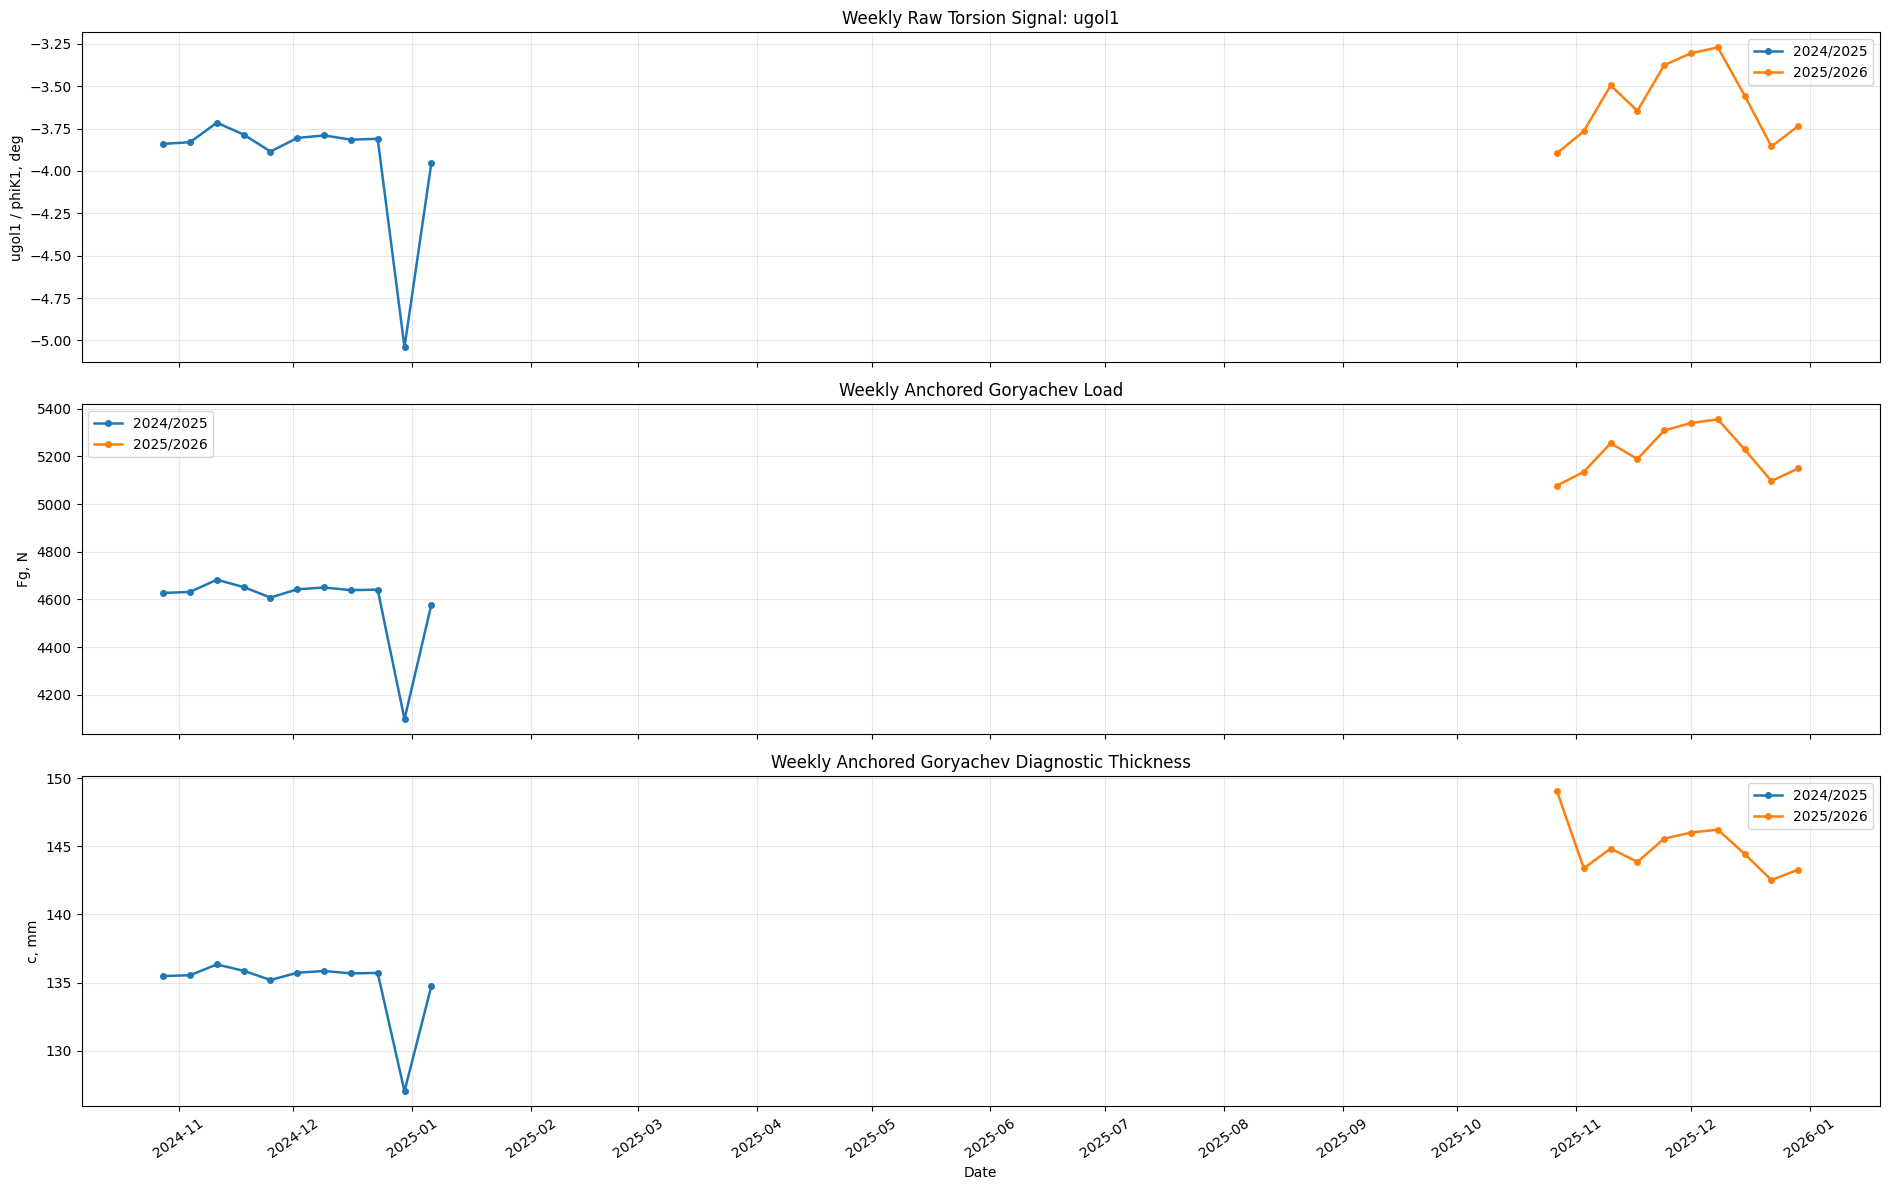

In [ ]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(19, 12),
    sharex=True,
)


for ice_season_year, group in weekly_raw_angle_summary.groupby(
    "iceSeasonStartYear"
):
    season_label = (
        f"{ice_season_year}/"
        f"{ice_season_year + 1}"
    )

    axes[0].plot(
        group["weekStart"],
        group["rawUgol1MedianDeg"],
        marker="o",
        linewidth=1.8,
        markersize=4,
        label=season_label,
    )

    axes[1].plot(
        group["weekStart"],
        group["FgMedianN"],
        marker="o",
        linewidth=1.8,
        markersize=4,
        label=season_label,
    )

    axes[2].plot(
        group["weekStart"],
        group["CmMedianMm"],
        marker="o",
        linewidth=1.8,
        markersize=4,
        label=season_label,
    )


axes[0].set_title(
    "Weekly Raw Torsion Signal: ugol1"
)

axes[0].set_ylabel(
    "ugol1 / phiK1, deg"
)

axes[1].set_title(
    "Weekly Anchored Goryachev Load"
)

axes[1].set_ylabel(
    "Fg, N"
)

axes[2].set_title(
    "Weekly Anchored Goryachev Diagnostic Thickness"
)

axes[2].set_ylabel(
    "c, mm"
)

axes[2].set_xlabel(
    "Date"
)


for axis in axes:
    axis.grid(
        True,
        alpha=0.30,
    )

    axis.legend(
        loc="best"
    )


axes[2].xaxis.set_major_locator(
    mdates.MonthLocator(
        interval=1
    )
)

axes[2].xaxis.set_major_formatter(
    mdates.DateFormatter(
        "%Y-%m"
    )
)

plt.xticks(
    rotation=35
)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd


assert "df_cal" in globals(), (
    "df_cal is unavailable."
)

assert "df_gor_raw_sensor_reference" in globals(), (
    "df_gor_raw_sensor_reference is unavailable. "
    "Run the raw sensor vs derived reference diagnostic first."
)


required_cal_columns = [
    "timestamp",
    "taC",
    "T1C",
    "vmpers",
    "currentA",
    "phiHdeg",
    "phiK1deg",
]

missing_cal_columns = [
    column
    for column in required_cal_columns
    if column not in df_cal.columns
]

assert not missing_cal_columns, (
    "df_cal is missing mechanical confounder columns: "
    f"{missing_cal_columns}"
)


df_gor_confounders = (
    df_gor_raw_sensor_reference[
        [
            "timestamp",
            "iceSeasonStartYear",
            "date",
            "winterPhase",
            "referenceKey",
            "deltaPhiHSensorDeg",
            "deltaPhiKSensorDeg",
            "deltaPhiKDeg",
            "gorFgAnchoredN",
            "gorCmAnchoredMm",
        ]
    ]
    .merge(
        df_cal[
            required_cal_columns
        ],
        on="timestamp",
        how="left",
        validate="one_to_one",
    )
    .copy()
)


for column in [
    "taC",
    "T1C",
    "vmpers",
    "currentA",
    "phiHdeg",
    "phiK1deg",
    "deltaPhiHSensorDeg",
    "deltaPhiKSensorDeg",
    "deltaPhiKDeg",
    "gorFgAnchoredN",
    "gorCmAnchoredMm",
]:
    df_gor_confounders[column] = pd.to_numeric(
        df_gor_confounders[column],
        errors="coerce",
    )


confounder_required_numeric = [
    "taC",
    "T1C",
    "vmpers",
    "currentA",
    "phiHdeg",
    "phiK1deg",
    "deltaPhiKSensorDeg",
    "gorFgAnchoredN",
    "gorCmAnchoredMm",
]

df_gor_confounders = (
    df_gor_confounders
    .dropna(
        subset=confounder_required_numeric
    )
    .sort_values(
        "timestamp"
    )
    .reset_index(
        drop=True
    )
)


daily_goryachev_confounders = (
    df_gor_confounders
    .groupby(
        [
            "iceSeasonStartYear",
            "date",
        ],
        as_index=False,
    )
    .agg(
        validRows=(
            "timestamp",
            "size",
        ),
        taC=(
            "taC",
            "median",
        ),
        T1C=(
            "T1C",
            "median",
        ),
        vmpers=(
            "vmpers",
            "median",
        ),
        currentA=(
            "currentA",
            "median",
        ),
        phiHdeg=(
            "phiHdeg",
            "median",
        ),
        phiK1deg=(
            "phiK1deg",
            "median",
        ),
        deltaPhiHSensorDeg=(
            "deltaPhiHSensorDeg",
            "median",
        ),
        deltaPhiKSensorDeg=(
            "deltaPhiKSensorDeg",
            "median",
        ),
        deltaPhiKDeg=(
            "deltaPhiKDeg",
            "median",
        ),
        gorFgAnchoredN=(
            "gorFgAnchoredN",
            "median",
        ),
        gorCmAnchoredMm=(
            "gorCmAnchoredMm",
            "median",
        ),
    )
    .sort_values(
        [
            "iceSeasonStartYear",
            "date",
        ]
    )
    .reset_index(
        drop=True
    )
)


correlation_rows = []

for ice_season_year, group in daily_goryachev_confounders.groupby(
    "iceSeasonStartYear"
):
    correlation_columns = [
        "taC",
        "T1C",
        "vmpers",
        "currentA",
        "phiHdeg",
        "deltaPhiHSensorDeg",
        "deltaPhiKSensorDeg",
        "gorFgAnchoredN",
        "gorCmAnchoredMm",
    ]

    correlation_matrix = (
        group[
            correlation_columns
        ]
        .corr(
            method="spearman"
        )
    )

    for response in [
        "deltaPhiKSensorDeg",
        "gorFgAnchoredN",
        "gorCmAnchoredMm",
    ]:
        for predictor in [
            "taC",
            "T1C",
            "vmpers",
            "currentA",
            "phiHdeg",
            "deltaPhiHSensorDeg",
        ]:
            correlation_rows.append(
                {
                    "iceSeason": (
                        f"{ice_season_year}/"
                        f"{ice_season_year + 1}"
                    ),
                    "response": response,
                    "predictor": predictor,
                    "spearmanCorrelation": (
                        correlation_matrix.loc[
                            response,
                            predictor,
                        ]
                    ),
                }
            )


df_gor_confounder_correlations = pd.DataFrame(
    correlation_rows
)


regression_rows = []

predictor_columns = [
    "taC",
    "T1C",
    "vmpers",
    "currentA",
    "phiHdeg",
]

for ice_season_year, group in daily_goryachev_confounders.groupby(
    "iceSeasonStartYear"
):
    regression_data = (
        group[
            predictor_columns
            + [
                "deltaPhiKSensorDeg",
            ]
        ]
        .dropna()
        .copy()
    )

    if len(regression_data) < 10:
        continue

    X_raw = regression_data[
        predictor_columns
    ].to_numpy(
        dtype=float
    )

    y_raw = regression_data[
        "deltaPhiKSensorDeg"
    ].to_numpy(
        dtype=float
    )

    X_mean = X_raw.mean(
        axis=0
    )

    X_std = X_raw.std(
        axis=0,
        ddof=0,
    )

    y_mean = y_raw.mean()

    y_std = y_raw.std(
        ddof=0
    )

    valid_predictors = (
        X_std > 0.0
    )

    X_standardized = (
        X_raw[
            :,
            valid_predictors,
        ]
        - X_mean[
            valid_predictors
        ]
    ) / X_std[
        valid_predictors
    ]

    y_standardized = (
        y_raw - y_mean
    ) / y_std

    X_design = np.column_stack(
        [
            np.ones(
                len(
                    X_standardized
                )
            ),
            X_standardized,
        ]
    )

    coefficients, residuals, rank, singular_values = np.linalg.lstsq(
        X_design,
        y_standardized,
        rcond=None,
    )

    y_predicted = (
        X_design
        @ coefficients
    )

    ss_total = np.sum(
        (
            y_standardized
            - y_standardized.mean()
        )
        ** 2
    )

    ss_residual = np.sum(
        (
            y_standardized
            - y_predicted
        )
        ** 2
    )

    r_squared = (
        1.0
        - ss_residual
        / ss_total
        if ss_total > 0.0
        else np.nan
    )

    active_predictors = np.array(
        predictor_columns
    )[
        valid_predictors
    ]

    for predictor, coefficient in zip(
        active_predictors,
        coefficients[1:],
    ):
        regression_rows.append(
            {
                "iceSeason": (
                    f"{ice_season_year}/"
                    f"{ice_season_year + 1}"
                ),
                "response": "deltaPhiKSensorDeg",
                "predictor": predictor,
                "standardizedCoefficient": coefficient,
                "modelR2": r_squared,
                "dailyPoints": len(
                    regression_data
                ),
            }
        )


df_gor_confounder_regression = pd.DataFrame(
    regression_rows
)


print("GORYACHEV MECHANICAL CONFOUNDER CORRELATIONS")
print("=" * 100)

display(
    df_gor_confounder_correlations
    .sort_values(
        [
            "iceSeason",
            "response",
            "spearmanCorrelation",
        ],
        ascending=[
            True,
            True,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)


print("\nSTANDARDIZED MODEL: DELTA PHIK SENSOR")
print("=" * 100)

display(
    df_gor_confounder_regression
    .sort_values(
        [
            "iceSeason",
            "standardizedCoefficient",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)


print("\nDAILY MECHANICAL-CONFOUNDER SIGNAL")
print("=" * 100)

display(
    daily_goryachev_confounders
)

GORYACHEV MECHANICAL CONFOUNDER CORRELATIONS


,iceSeason,response,predictor,spearmanCorrelation
0,2024/2025,deltaPhiKSensorDeg,phiHdeg,0.235216
1,2024/2025,deltaPhiKSensorDeg,deltaPhiHSensorDeg,0.235216
2,2024/2025,deltaPhiKSensorDeg,currentA,0.113141
3,2024/2025,deltaPhiKSensorDeg,taC,-0.125800
4,2024/2025,deltaPhiKSensorDeg,T1C,-0.132161
5,2024/2025,deltaPhiKSensorDeg,vmpers,NaN
6,2024/2025,gorCmAnchoredMm,phiHdeg,0.231365
7,2024/2025,gorCmAnchoredMm,deltaPhiHSensorDeg,0.231365
8,2024/2025,gorCmAnchoredMm,currentA,0.091410
9,2024/2025,gorCmAnchoredMm,taC,-0.148482



STANDARDIZED MODEL: DELTA PHIK SENSOR


,iceSeason,response,predictor,standardizedCoefficient,modelR2,dailyPoints
0,2024/2025,deltaPhiKSensorDeg,taC,2.991385,0.107285,58
1,2024/2025,deltaPhiKSensorDeg,phiHdeg,0.222891,0.107285,58
2,2024/2025,deltaPhiKSensorDeg,currentA,-0.052887,0.107285,58
3,2024/2025,deltaPhiKSensorDeg,T1C,-2.879404,0.107285,58
4,2025/2026,deltaPhiKSensorDeg,T1C,7.580421,0.162566,62
5,2025/2026,deltaPhiKSensorDeg,currentA,0.155388,0.162566,62
6,2025/2026,deltaPhiKSensorDeg,phiHdeg,-0.030314,0.162566,62
7,2025/2026,deltaPhiKSensorDeg,vmpers,-0.142191,0.162566,62
8,2025/2026,deltaPhiKSensorDeg,taC,-7.645871,0.162566,62



DAILY MECHANICAL-CONFOUNDER SIGNAL


,iceSeasonStartYear,date,validRows,taC,T1C,vmpers,currentA,phiHdeg,phiK1deg,deltaPhiHSensorDeg,deltaPhiKSensorDeg,deltaPhiKDeg,gorFgAnchoredN,gorCmAnchoredMm
0,2024,2024-11-01,6,-17.80,-15.7,0.0,23.0,2.445,-3.890,-0.080,-0.055,10.421095,4604.742011,135.132203
1,2024,2024-11-02,9,-20.80,-18.6,0.0,24.0,2.495,-3.785,-0.030,0.050,10.526095,4651.421291,135.847305
2,2024,2024-11-03,7,-21.50,-19.9,0.0,28.0,2.625,-3.805,0.100,0.030,10.506095,4642.855707,135.718348
3,2024,2024-11-04,9,-21.30,-19.0,0.0,27.0,2.565,-3.745,0.040,0.090,10.566095,4669.233759,136.117769
4,2024,2024-11-05,4,-29.45,-27.1,0.0,27.5,2.750,-3.430,0.225,0.405,10.881095,4809.403891,138.238276
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,2025,2025-12-28,134,-43.40,-40.7,0.0,23.0,2.530,-3.785,0.175,0.370,11.600714,5127.885614,142.969429
116,2025,2025-12-29,137,-41.80,-39.3,0.0,28.0,2.265,-3.425,-0.090,0.730,11.960714,5286.457922,145.243994
117,2025,2025-12-30,134,-43.45,-40.9,0.0,28.0,2.525,-3.790,0.170,0.365,11.595714,5125.674576,142.937209
118,2025,2025-12-31,133,-44.10,-41.4,0.0,29.0,2.575,-3.855,0.220,0.300,11.530714,5097.045006,142.522787


In [ ]:
import math
import numpy as np
import pandas as pd

from src.goryachev_model import (
    eq6_tension,
    eq12_ice_wall_thickness,
)


assert "df_gor_l0t_anchor" in globals(), (
    "df_gor_l0t_anchor is unavailable."
)

assert "cable_params" in globals(), (
    "cable_params is unavailable."
)


def get_cable_parameter(
    parameter_object,
    candidates: list[str],
    semantic_name: str,
) -> float:
    for attribute_name in candidates:
        if hasattr(
            parameter_object,
            attribute_name,
        ):
            value = getattr(
                parameter_object,
                attribute_name,
            )

            if value is not None:
                return float(value)

    raise AttributeError(
        f"Cannot resolve {semantic_name}. "
        f"Candidates: {candidates}"
    )


CABLE_L_M = get_cable_parameter(
    parameter_object=cable_params,
    candidates=[
        "lm",
        "lM",
        "L_M",
    ],
    semantic_name="span length",
)

CABLE_B_N_M2 = get_cable_parameter(
    parameter_object=cable_params,
    candidates=[
        "BNm2",
        "bNm2",
        "B_N_M2",
    ],
    semantic_name="B",
)

CABLE_C_N_M = get_cable_parameter(
    parameter_object=cable_params,
    candidates=[
        "CNm",
        "cNm",
        "C_N_M",
    ],
    semantic_name="C",
)

CABLE_D_PR_M = get_cable_parameter(
    parameter_object=cable_params,
    candidates=[
        "dprm",
        "dPrM",
        "D_PR_M",
    ],
    semantic_name="bare conductor diameter",
)


required_columns = [
    "timestamp",
    "gorL0gAnchorStatus",
    "phiHdeg",
    "phiK1deg",
    "referencePhiK0Rad",
    "referenceAlphaStarPerN",
    "gorL0gAnchoredM",
    "rhotkgm3",
    "gorFgAnchoredN",
    "gorCmAnchoredMm",
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_gor_l0t_anchor.columns
]

assert not missing_columns, (
    "Missing columns: "
    f"{missing_columns}"
)


df_gor_sensitivity = (
    df_gor_l0t_anchor
    .loc[
        df_gor_l0t_anchor[
            "gorL0gAnchorStatus"
        ]
        .eq("ok"),
        required_columns,
    ]
    .copy()
)


df_gor_sensitivity["timestamp"] = pd.to_datetime(
    df_gor_sensitivity["timestamp"],
    errors="coerce",
)

df_gor_sensitivity = (
    df_gor_sensitivity
    .dropna(
        subset=[
            "timestamp",
            "phiHdeg",
            "phiK1deg",
            "referencePhiK0Rad",
            "referenceAlphaStarPerN",
            "gorL0gAnchoredM",
            "rhotkgm3",
        ]
    )
    .copy()
)


df_gor_sensitivity["month"] = (
    df_gor_sensitivity[
        "timestamp"
    ]
    .dt.month
)

df_gor_sensitivity = (
    df_gor_sensitivity
    .loc[
        df_gor_sensitivity[
            "month"
        ]
        .isin(
            [
                11,
                12,
                1,
                2,
            ]
        )
    ]
    .copy()
)


SENSITIVITY_STEP_DEG = 0.01

df_gor_sensitivity[
    "dFg_dPhiK_N_per_deg"
] = np.nan

df_gor_sensitivity[
    "dFg_dPhiH_N_per_deg"
] = np.nan

df_gor_sensitivity[
    "dCm_dPhiK_mm_per_deg"
] = np.nan

df_gor_sensitivity[
    "dCm_dPhiH_mm_per_deg"
] = np.nan

df_gor_sensitivity[
    "sensitivityStatus"
] = "not_calculated"


def calculate_fg_and_cm(
    phiH_deg: float,
    phiK1_deg: float,
    phiK0_rad: float,
    alpha_star: float,
    L0g_m: float,
    rho_kg_m3: float,
) -> tuple[float, float]:
    fg_n = eq6_tension(
        phiH_deg=float(
            phiH_deg
        ),
        phiK1_rad=math.radians(
            float(
                phiK1_deg
            )
        ),
        phiK0_rad=float(
            phiK0_rad
        ),
        alpha_star=float(
            alpha_star
        ),
        L0g=float(
            L0g_m
        ),
        l=CABLE_L_M,
        B=CABLE_B_N_M2,
        C=CABLE_C_N_M,
    )

    cm_m = eq12_ice_wall_thickness(
        d_pr=CABLE_D_PR_M,
        Fg=float(
            fg_n
        ),
        q0g=float(
            rho_kg_m3
        ),
        L0g=float(
            L0g_m
        ),
    )

    return (
        float(
            fg_n
        ),
        float(
            cm_m
        ) * 1000.0,
    )


for row_index in df_gor_sensitivity.index:
    row = df_gor_sensitivity.loc[
        row_index
    ]

    try:
        base_fg, base_cm = calculate_fg_and_cm(
            phiH_deg=float(
                row["phiHdeg"]
            ),
            phiK1_deg=float(
                row["phiK1deg"]
            ),
            phiK0_rad=float(
                row[
                    "referencePhiK0Rad"
                ]
            ),
            alpha_star=float(
                row[
                    "referenceAlphaStarPerN"
                ]
            ),
            L0g_m=float(
                row[
                    "gorL0gAnchoredM"
                ]
            ),
            rho_kg_m3=float(
                row[
                    "rhotkgm3"
                ]
            ),
        )

        fg_k_plus, cm_k_plus = calculate_fg_and_cm(
            phiH_deg=float(
                row["phiHdeg"]
            ),
            phiK1_deg=float(
                row["phiK1deg"]
            )
            + SENSITIVITY_STEP_DEG,
            phiK0_rad=float(
                row[
                    "referencePhiK0Rad"
                ]
            ),
            alpha_star=float(
                row[
                    "referenceAlphaStarPerN"
                ]
            ),
            L0g_m=float(
                row[
                    "gorL0gAnchoredM"
                ]
            ),
            rho_kg_m3=float(
                row[
                    "rhotkgm3"
                ]
            ),
        )

        fg_k_minus, cm_k_minus = calculate_fg_and_cm(
            phiH_deg=float(
                row["phiHdeg"]
            ),
            phiK1_deg=float(
                row["phiK1deg"]
            )
            - SENSITIVITY_STEP_DEG,
            phiK0_rad=float(
                row[
                    "referencePhiK0Rad"
                ]
            ),
            alpha_star=float(
                row[
                    "referenceAlphaStarPerN"
                ]
            ),
            L0g_m=float(
                row[
                    "gorL0gAnchoredM"
                ]
            ),
            rho_kg_m3=float(
                row[
                    "rhotkgm3"
                ]
            ),
        )

        fg_h_plus, cm_h_plus = calculate_fg_and_cm(
            phiH_deg=float(
                row["phiHdeg"]
            )
            + SENSITIVITY_STEP_DEG,
            phiK1_deg=float(
                row["phiK1deg"]
            ),
            phiK0_rad=float(
                row[
                    "referencePhiK0Rad"
                ]
            ),
            alpha_star=float(
                row[
                    "referenceAlphaStarPerN"
                ]
            ),
            L0g_m=float(
                row[
                    "gorL0gAnchoredM"
                ]
            ),
            rho_kg_m3=float(
                row[
                    "rhotkgm3"
                ]
            ),
        )

        fg_h_minus, cm_h_minus = calculate_fg_and_cm(
            phiH_deg=float(
                row["phiHdeg"]
            )
            - SENSITIVITY_STEP_DEG,
            phiK1_deg=float(
                row["phiK1deg"]
            ),
            phiK0_rad=float(
                row[
                    "referencePhiK0Rad"
                ]
            ),
            alpha_star=float(
                row[
                    "referenceAlphaStarPerN"
                ]
            ),
            L0g_m=float(
                row[
                    "gorL0gAnchoredM"
                ]
            ),
            rho_kg_m3=float(
                row[
                    "rhotkgm3"
                ]
            ),
        )

        df_gor_sensitivity.loc[
            row_index,
            "dFg_dPhiK_N_per_deg",
        ] = (
            fg_k_plus
            - fg_k_minus
        ) / (
            2.0
            * SENSITIVITY_STEP_DEG
        )

        df_gor_sensitivity.loc[
            row_index,
            "dFg_dPhiH_N_per_deg",
        ] = (
            fg_h_plus
            - fg_h_minus
        ) / (
            2.0
            * SENSITIVITY_STEP_DEG
        )

        df_gor_sensitivity.loc[
            row_index,
            "dCm_dPhiK_mm_per_deg",
        ] = (
            cm_k_plus
            - cm_k_minus
        ) / (
            2.0
            * SENSITIVITY_STEP_DEG
        )

        df_gor_sensitivity.loc[
            row_index,
            "dCm_dPhiH_mm_per_deg",
        ] = (
            cm_h_plus
            - cm_h_minus
        ) / (
            2.0
            * SENSITIVITY_STEP_DEG
        )

        df_gor_sensitivity.loc[
            row_index,
            "sensitivityStatus",
        ] = "ok"

    except Exception as exc:
        df_gor_sensitivity.loc[
            row_index,
            "sensitivityStatus",
        ] = (
            f"error_{type(exc).__name__}"
        )


df_gor_sensitivity_ok = (
    df_gor_sensitivity
    .loc[
        df_gor_sensitivity[
            "sensitivityStatus"
        ]
        .eq("ok")
    ]
    .copy()
)


df_gor_sensitivity_ok[
    "absSensitivityRatioKtoH_Fg"
] = (
    df_gor_sensitivity_ok[
        "dFg_dPhiK_N_per_deg"
    ]
    .abs()
    / df_gor_sensitivity_ok[
        "dFg_dPhiH_N_per_deg"
    ]
    .abs()
    .replace(
        0.0,
        np.nan,
    )
)

df_gor_sensitivity_ok[
    "absSensitivityRatioKtoH_Cm"
] = (
    df_gor_sensitivity_ok[
        "dCm_dPhiK_mm_per_deg"
    ]
    .abs()
    / df_gor_sensitivity_ok[
        "dCm_dPhiH_mm_per_deg"
    ]
    .abs()
    .replace(
        0.0,
        np.nan,
    )
)


df_gor_sensitivity_ok[
    "iceSeason"
] = np.where(
    df_gor_sensitivity_ok[
        "timestamp"
    ]
    .dt.month
    .ge(11),
    (
        df_gor_sensitivity_ok[
            "timestamp"
        ]
        .dt.year.astype(str)
        + "/"
        + (
            df_gor_sensitivity_ok[
                "timestamp"
            ]
            .dt.year
            + 1
        )
        .astype(str)
    ),
    (
        (
            df_gor_sensitivity_ok[
                "timestamp"
            ]
            .dt.year
            - 1
        )
        .astype(str)
        + "/"
        + df_gor_sensitivity_ok[
            "timestamp"
        ]
        .dt.year.astype(str)
    ),
)


sensitivity_summary = (
    df_gor_sensitivity_ok
    .groupby(
        "iceSeason",
        as_index=False,
    )
    .agg(
        validRows=(
            "timestamp",
            "size",
        ),
        median_dFg_dPhiK_N_per_deg=(
            "dFg_dPhiK_N_per_deg",
            "median",
        ),
        median_dFg_dPhiH_N_per_deg=(
            "dFg_dPhiH_N_per_deg",
            "median",
        ),
        median_dCm_dPhiK_mm_per_deg=(
            "dCm_dPhiK_mm_per_deg",
            "median",
        ),
        median_dCm_dPhiH_mm_per_deg=(
            "dCm_dPhiH_mm_per_deg",
            "median",
        ),
        medianAbsRatioKtoH_Fg=(
            "absSensitivityRatioKtoH_Fg",
            "median",
        ),
        medianAbsRatioKtoH_Cm=(
            "absSensitivityRatioKtoH_Cm",
            "median",
        ),
        p95AbsRatioKtoH_Cm=(
            "absSensitivityRatioKtoH_Cm",
            lambda series: series.quantile(
                0.95
            ),
        ),
    )
)


print("GORYACHEV LOCAL SENSITIVITY SUMMARY")
print("=" * 100)

display(
    sensitivity_summary
)


print("\nSENSITIVITY STATUS COUNTS")
print("=" * 100)

display(
    df_gor_sensitivity[
        "sensitivityStatus"
    ]
    .value_counts(
        dropna=False
    )
    .rename(
        "count"
    )
    .to_frame()
)

GORYACHEV LOCAL SENSITIVITY SUMMARY


,iceSeason,validRows,median_dFg_dPhiK_N_per_deg,median_dFg_dPhiH_N_per_deg,median_dCm_dPhiK_mm_per_deg,median_dCm_dPhiH_mm_per_deg,medianAbsRatioKtoH_Fg,medianAbsRatioKtoH_Cm,p95AbsRatioKtoH_Cm
0,2024/2025,404,442.088770,1.796351,6.723872,0.027334,246.108253,246.108281,279.005293
1,2025/2026,7673,442.198748,2.116821,6.335988,0.030571,208.861626,208.861647,238.868905



SENSITIVITY STATUS COUNTS


,count
sensitivityStatus,
ok,8077


In [ ]:
import pandas as pd


assert "df_cal" in globals(), (
    "df_cal is unavailable."
)

assert "df_sim" in globals(), (
    "df_sim is unavailable."
)

assert "df_goryachev_reference_states" in globals(), (
    "df_goryachev_reference_states is unavailable."
)


def find_related_columns(
    dataframe: pd.DataFrame,
    tokens: list[str],
) -> list[str]:
    return [
        column
        for column in dataframe.columns
        if any(
            token.lower()
            in column.lower()
            for token in tokens
        )
    ]


print("DF_CAL REFERENCE-RELATED COLUMNS")
print("=" * 100)

print(
    find_related_columns(
        dataframe=df_cal,
        tokens=[
            "reference",
            "orientation",
            "segment",
            "month",
            "noice",
            "angle",
            "ugol",
            "phi",
        ],
    )
)


print("\nDF_SIM REFERENCE-RELATED COLUMNS")
print("=" * 100)

print(
    find_related_columns(
        dataframe=df_sim,
        tokens=[
            "reference",
            "orientation",
            "segment",
            "month",
            "gor",
        ],
    )
)


print("\nREFERENCE-STATE TABLE COLUMNS")
print("=" * 100)

print(
    df_goryachev_reference_states.columns.tolist()
)


print("\nDF_CAL: NO-ICE REFERENCE COUNTS")
print("=" * 100)

if "isNoIceReference" in df_cal.columns:
    display(
        df_cal[
            "isNoIceReference"
        ]
        .value_counts(
            dropna=False,
        )
        .rename(
            "count"
        )
        .to_frame()
    )
else:
    print(
        "isNoIceReference is absent from df_cal."
    )


print("\nREFERENCE-STATE TABLE")
print("=" * 100)

display(
    df_goryachev_reference_states
)


print("\nDF_CAL SAMPLE WITH RAW ANGLES")
print("=" * 100)

candidate_columns = [
    column
    for column in [
        "timestamp",
        "isNoIceReference",
        "ugol1DegRaw",
        "ugol2DegRaw",
        "phiHdeg",
        "phiK1deg",
        "orientationSegmentId",
        "orientationReferenceMonth",
        "orientationReferenceKey",
        "orientationBaselineAvailable",
        "anglesValidForGoryachev",
    ]
    if column in df_cal.columns
]

display(
    df_cal[
        candidate_columns
    ]
    .head(20)
)


print("\nDF_SIM SAMPLE WITH GORYACHEV REFERENCE FIELDS")
print("=" * 100)

candidate_columns = [
    column
    for column in [
        "timestamp",
        "gorStatus",
        "gorReferenceKey",
        "gorReferenceSegmentId",
        "orientationReferenceKey",
        "orientationSegmentId",
        "rhotkgm3",
        "gorFgN",
        "gorCm",
    ]
    if column in df_sim.columns
]

display(
    df_sim[
        candidate_columns
    ]
    .head(20)
)

DF_CAL REFERENCE-RELATED COLUMNS
['phiHdeg', 'phiK1deg', 'isNoIceReference', 'ugol1DegRaw', 'ugol2DegRaw', 'rawAnglesAvailable', 'rawAngleSource', 'rawAngleFieldsVersion', 'phiHdegRawValid', 'phiK1degRawValid', 'anglesValidForGoryachev', 'rawPhiHSource', 'rawPhiK1Source', 'angleMapping', 'rawAngleValid', 'rawAngleSegmentId', 'rawAngleSegmentStart', 'rawAngleSegmentReason', 'rawAngleChangeDetected', 'rawAngleChangeMagnitudeUgol1Deg', 'rawAngleChangeMagnitudeUgol2Deg', 'rawAngleSegmentValid', 'orientationSegmentId', 'canonicalAngleSegmentId', 'canonicalAngleSegmentRole', 'rawAngleMacroSegmentId', 'canonicalAngleSegmentationMode', 'isAngleTransition', 'isEligibleForGoryachevReference', 'thermalNoIceReference', 'seasonalNoIceReference', 'isGoryachevReferenceCandidate', 'goryachevReferenceSource', 'orientationMonth', 'orientationMonthStr', 'orientationReferenceKey', 'orientationReferenceMonth', 'orientationAssignmentMode', 'orientationBaselineUgol1Deg', 'orientationBaselineUgol2Deg', 'orien

,count
isNoIceReference,
False,36669
True,19725



REFERENCE-STATE TABLE


,orientationSegmentId,nReferenceRows,TcalC,phiHcalDeg,phiK1calDeg,phiK0calDeg,alphaStarPerN,q0CalNPerM,L0CalM,L0TCalM,L0gCalM,FgCalN,SagCalM,phiK1calRad,phiK0calRad,orientationReferenceMonth,goryachevReferenceKey
0,1.0,237,-12.8,2.585,-3.745,-13.980582,1.526795e-07,2.701701,150.947143,151.042263,150.947143,4522.499683,1.704025,-0.065363,-0.244007,2024-03,1|2024-03
1,1.0,217,-0.4,2.535,-3.835,-14.268323,1.526795e-07,2.701058,150.943153,151.002298,150.943153,4609.871255,1.671033,-0.066933,-0.249029,2024-04,1|2024-04
2,1.0,229,10.1,2.545,-3.820,-14.209271,1.526795e-07,2.700513,150.943981,150.972678,150.943981,4590.405874,1.677631,-0.066672,-0.247999,2024-05,1|2024-05
3,1.0,216,20.9,2.540,-3.815,-14.221446,1.526795e-07,2.699953,150.943600,150.940991,150.943600,4597.993932,1.674332,-0.066584,-0.248211,2024-06,1|2024-06
4,1.0,50,23.1,2.545,-3.815,-14.200386,1.526795e-07,2.699839,150.944007,150.935023,150.944007,4588.688042,1.677631,-0.066584,-0.247843,2024-07,1|2024-07
5,1.0,22,12.7,2.560,-3.760,-14.087748,1.526795e-07,2.700378,150.945192,150.966351,150.945192,4563.221526,1.687529,-0.065624,-0.245878,2024-08,1|2024-08
6,1.0,248,6.3,2.545,-3.815,-14.205407,1.526795e-07,2.700710,150.943973,150.983688,150.943973,4590.908226,1.677631,-0.066584,-0.247931,2024-09,1|2024-09
7,1.0,243,-5.5,2.525,-3.835,-14.311095,1.526795e-07,2.701323,150.942335,151.016272,150.942335,4628.771420,1.664435,-0.066933,-0.249776,2024-10,1|2024-10
8,3.0,4541,-17.7,2.525,-3.725,-14.204776,1.526795e-07,2.701956,150.942310,151.051647,150.942310,4630.398618,1.664435,-0.065014,-0.247920,2025-03,3|2025-03
9,3.0,3647,2.6,2.485,-3.915,-14.556893,1.526795e-07,2.700902,150.939101,150.989544,150.939101,4702.032515,1.638042,-0.068330,-0.254066,2025-04,3|2025-04



DF_CAL SAMPLE WITH RAW ANGLES


,timestamp,isNoIceReference,ugol1DegRaw,ugol2DegRaw,phiHdeg,phiK1deg,orientationSegmentId,orientationReferenceMonth,orientationReferenceKey,orientationBaselineAvailable,anglesValidForGoryachev
0,2023-10-19 01:22:36,True,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,False,False
1,2023-10-19 01:33:08,True,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,False,False
2,2023-12-13 05:43:48,False,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,False,False
3,2023-12-13 09:02:46,False,-3.645,-2.305,2.305,-3.645,1,<NA>,<NA>,False,True
4,2023-12-13 12:21:47,False,-3.685,-2.315,2.315,-3.685,1,<NA>,<NA>,False,True
5,2023-12-13 15:40:47,False,-3.685,-2.315,2.315,-3.685,1,<NA>,<NA>,False,True
6,2023-12-13 18:59:45,False,-3.675,-2.395,2.395,-3.675,1,<NA>,<NA>,False,True
7,2023-12-13 22:19:08,False,-3.815,-2.725,2.725,-3.815,1,<NA>,<NA>,False,True
8,2023-12-14 01:38:41,False,-3.855,-2.785,2.785,-3.855,1,<NA>,<NA>,False,True
9,2023-12-14 04:58:12,False,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,False,False



DF_SIM SAMPLE WITH GORYACHEV REFERENCE FIELDS


,timestamp,gorStatus,gorReferenceKey,gorReferenceSegmentId,orientationReferenceKey,orientationSegmentId,rhotkgm3,gorFgN,gorCm
0,2023-10-19 01:22:36,no_ice,<NA>,NaN,<NA>,NaN,0.0,NaN,0.0
1,2023-10-19 01:33:08,no_ice,<NA>,NaN,<NA>,NaN,0.0,NaN,0.0
2,2023-12-13 05:43:48,angle_out_of_range,<NA>,NaN,<NA>,NaN,50.0,NaN,NaN
3,2023-12-13 09:02:46,no_reference_for_raw_angle_segment,<NA>,NaN,<NA>,NaN,50.0,NaN,NaN
4,2023-12-13 12:21:47,no_reference_for_raw_angle_segment,<NA>,NaN,<NA>,NaN,50.0,NaN,NaN
5,2023-12-13 15:40:47,no_reference_for_raw_angle_segment,<NA>,NaN,<NA>,NaN,50.0,NaN,NaN
6,2023-12-13 18:59:45,no_reference_for_raw_angle_segment,<NA>,NaN,<NA>,NaN,50.0,NaN,NaN
7,2023-12-13 22:19:08,no_reference_for_raw_angle_segment,<NA>,NaN,<NA>,NaN,50.0,NaN,NaN
8,2023-12-14 01:38:41,no_reference_for_raw_angle_segment,<NA>,NaN,<NA>,NaN,50.0,NaN,NaN
9,2023-12-14 04:58:12,angle_out_of_range,<NA>,NaN,<NA>,NaN,50.0,NaN,NaN


In [ ]:
import math
import numpy as np
import pandas as pd

from src.goryachev_model import (
    eq1_q0_from_temperature,
    eq2_L0,
    eq3_L0T,
    eq4_phiK0_rad,
    eq5_L0g,
    eq6_tension,
    eq12_ice_wall_thickness,
)


assert "df_cal" in globals(), (
    "df_cal is unavailable."
)

assert "df_sim" in globals(), (
    "df_sim is unavailable."
)

assert "cable_params" in globals(), (
    "cable_params is unavailable."
)


def get_cable_parameter(
    parameter_object,
    candidates: list[str],
    semantic_name: str,
) -> float:
    for attribute_name in candidates:
        if hasattr(
            parameter_object,
            attribute_name,
        ):
            value = getattr(
                parameter_object,
                attribute_name,
            )

            if value is not None:
                return float(value)

    raise AttributeError(
        f"Cannot resolve cable parameter: "
        f"{semantic_name}. "
        f"Candidates: {candidates}"
    )


def safe_float(
    value,
) -> float:
    try:
        numeric_value = float(value)

        if math.isfinite(
            numeric_value
        ):
            return numeric_value

    except (
        TypeError,
        ValueError,
    ):
        pass

    return np.nan


CABLE_L_M = get_cable_parameter(
    parameter_object=cable_params,
    candidates=[
        "lm",
        "lM",
        "L_M",
    ],
    semantic_name="span length",
)

CABLE_B_N_M2 = get_cable_parameter(
    parameter_object=cable_params,
    candidates=[
        "BNm2",
        "bNm2",
        "B_N_M2",
    ],
    semantic_name="B",
)

CABLE_C_N_M = get_cable_parameter(
    parameter_object=cable_params,
    candidates=[
        "CNm",
        "cNm",
        "C_N_M",
    ],
    semantic_name="C",
)

CABLE_D_PR_M = get_cable_parameter(
    parameter_object=cable_params,
    candidates=[
        "dprm",
        "dPrM",
        "D_PR_M",
    ],
    semantic_name="bare conductor diameter",
)

CABLE_Q0T_N_PER_M = get_cable_parameter(
    parameter_object=cable_params,
    candidates=[
        "q0TNperm",
        "q0TNPerM",
        "q0tNperm",
        "q0tNPerM",
    ],
    semantic_name="q0T",
)

CABLE_BETA_1_PER_C = get_cable_parameter(
    parameter_object=cable_params,
    candidates=[
        "beta1perC",
        "beta1PerC",
    ],
    semantic_name="beta",
)

CABLE_T0_C = get_cable_parameter(
    parameter_object=cable_params,
    candidates=[
        "T0C",
        "t0C",
    ],
    semantic_name="T0",
)


CABLE_ALPHA_STAR_PER_N = 1.0 / (
    get_cable_parameter(
        parameter_object=cable_params,
        candidates=[
            "AN",
            "aN",
            "A_N",
        ],
        semantic_name="A",
    )
    - (
        CABLE_C_N_M
        ** 2
        / CABLE_B_N_M2
    )
)


required_cal_columns = [
    "timestamp",
    "T1C",
    "ugol1DegRaw",
    "ugol2DegRaw",
    "isGoryachevReferenceCandidate",
    "orientationReferenceKey",
    "anglesValidForGoryachev",
]

missing_cal_columns = [
    column
    for column in required_cal_columns
    if column not in df_cal.columns
]

assert not missing_cal_columns, (
    "df_cal is missing columns: "
    f"{missing_cal_columns}"
)


required_sim_columns = [
    "timestamp",
    "gorStatus",
    "gorReferenceKey",
    "rhotkgm3",
]

missing_sim_columns = [
    column
    for column in required_sim_columns
    if column not in df_sim.columns
]

assert not missing_sim_columns, (
    "df_sim is missing columns: "
    f"{missing_sim_columns}"
)


df_mapping_cal = (
    df_cal[
        required_cal_columns
    ]
    .copy()
)

df_mapping_cal["timestamp"] = pd.to_datetime(
    df_mapping_cal["timestamp"],
    errors="coerce",
)

df_mapping_cal = (
    df_mapping_cal
    .dropna(
        subset=[
            "timestamp",
        ]
    )
    .sort_values(
        "timestamp"
    )
    .reset_index(
        drop=True
    )
)


for column in [
    "T1C",
    "ugol1DegRaw",
    "ugol2DegRaw",
]:
    df_mapping_cal[column] = pd.to_numeric(
        df_mapping_cal[column],
        errors="coerce",
    )


df_mapping_cal[
    "isGoryachevReferenceCandidate"
] = (
    df_mapping_cal[
        "isGoryachevReferenceCandidate"
    ]
    .fillna(False)
    .astype(bool)
)

df_mapping_cal[
    "anglesValidForGoryachev"
] = (
    df_mapping_cal[
        "anglesValidForGoryachev"
    ]
    .fillna(False)
    .astype(bool)
)


df_mapping_sim = (
    df_sim[
        required_sim_columns
    ]
    .copy()
)

df_mapping_sim["timestamp"] = pd.to_datetime(
    df_mapping_sim["timestamp"],
    errors="coerce",
)

df_mapping_sim = (
    df_mapping_sim
    .dropna(
        subset=[
            "timestamp",
        ]
    )
    .sort_values(
        "timestamp"
    )
    .drop_duplicates(
        subset=[
            "timestamp",
        ],
        keep="last",
    )
    .reset_index(
        drop=True
    )
)

df_mapping_sim["rhotkgm3"] = pd.to_numeric(
    df_mapping_sim["rhotkgm3"],
    errors="coerce",
)


df_mapping_runtime = (
    df_mapping_cal
    .merge(
        df_mapping_sim,
        on="timestamp",
        how="inner",
        validate="one_to_one",
    )
    .copy()
)


df_mapping_reference_candidates = (
    df_mapping_cal
    .loc[
        df_mapping_cal[
            "isGoryachevReferenceCandidate"
        ]
        & df_mapping_cal[
            "anglesValidForGoryachev"
        ]
        & df_mapping_cal[
            "orientationReferenceKey"
        ]
        .notna()
        & df_mapping_cal[
            "T1C"
        ]
        .notna()
        & df_mapping_cal[
            "ugol1DegRaw"
        ]
        .notna()
        & df_mapping_cal[
            "ugol2DegRaw"
        ]
        .notna()
    ]
    .copy()
)


df_mapping_runtime = (
    df_mapping_runtime
    .loc[
        df_mapping_runtime[
            "gorStatus"
        ]
        .eq("ok")
        & df_mapping_runtime[
            "gorReferenceKey"
        ]
        .notna()
        & df_mapping_runtime[
            "T1C"
        ]
        .notna()
        & df_mapping_runtime[
            "ugol1DegRaw"
        ]
        .notna()
        & df_mapping_runtime[
            "ugol2DegRaw"
        ]
        .notna()
        & df_mapping_runtime[
            "rhotkgm3"
        ]
        .gt(0.0)
    ]
    .copy()
)


print("CANDIDATE-MAPPING INPUT SIZES")
print("=" * 100)

print(
    "Reference candidate rows:",
    len(df_mapping_reference_candidates),
)

print(
    "Reference keys:",
    df_mapping_reference_candidates[
        "orientationReferenceKey"
    ]
    .nunique(),
)

print(
    "Current valid Goryachev runtime rows:",
    len(df_mapping_runtime),
)

print(
    "Current runtime reference keys:",
    df_mapping_runtime[
        "gorReferenceKey"
    ]
    .nunique(),
)


MAPPING_CANDIDATES = [
    {
        "mappingId": "M1_current_phiH_negU2_phiK_posU1",
        "phiHSource": "ugol2DegRaw",
        "phiHSign": -1.0,
        "phiKSource": "ugol1DegRaw",
        "phiKSign": +1.0,
    },
    {
        "mappingId": "M2_phiH_posU2_phiK_posU1",
        "phiHSource": "ugol2DegRaw",
        "phiHSign": +1.0,
        "phiKSource": "ugol1DegRaw",
        "phiKSign": +1.0,
    },
    {
        "mappingId": "M3_phiH_negU2_phiK_negU1",
        "phiHSource": "ugol2DegRaw",
        "phiHSign": -1.0,
        "phiKSource": "ugol1DegRaw",
        "phiKSign": -1.0,
    },
    {
        "mappingId": "M4_phiH_posU2_phiK_negU1",
        "phiHSource": "ugol2DegRaw",
        "phiHSign": +1.0,
        "phiKSource": "ugol1DegRaw",
        "phiKSign": -1.0,
    },
    {
        "mappingId": "M5_swapped_phiH_negU1_phiK_posU2",
        "phiHSource": "ugol1DegRaw",
        "phiHSign": -1.0,
        "phiKSource": "ugol2DegRaw",
        "phiKSign": +1.0,
    },
    {
        "mappingId": "M6_swapped_phiH_posU1_phiK_posU2",
        "phiHSource": "ugol1DegRaw",
        "phiHSign": +1.0,
        "phiKSource": "ugol2DegRaw",
        "phiKSign": +1.0,
    },
    {
        "mappingId": "M7_swapped_phiH_negU1_phiK_negU2",
        "phiHSource": "ugol1DegRaw",
        "phiHSign": -1.0,
        "phiKSource": "ugol2DegRaw",
        "phiKSign": -1.0,
    },
    {
        "mappingId": "M8_swapped_phiH_posU1_phiK_negU2",
        "phiHSource": "ugol1DegRaw",
        "phiHSign": +1.0,
        "phiKSource": "ugol2DegRaw",
        "phiKSign": -1.0,
    },
]


def add_candidate_angles(
    dataframe: pd.DataFrame,
    mapping: dict,
) -> pd.DataFrame:
    result = dataframe.copy()

    result["candidatePhiHdeg"] = (
        float(
            mapping["phiHSign"]
        )
        * result[
            mapping["phiHSource"]
        ]
    )

    result["candidatePhiK1deg"] = (
        float(
            mapping["phiKSign"]
        )
        * result[
            mapping["phiKSource"]
        ]
    )

    return result


def build_reference_state(
    reference_rows: pd.DataFrame,
) -> dict:
    if len(reference_rows) < 5:
        return {
            "status": "insufficient_reference_rows",
        }

    t_cal_c = safe_float(
        reference_rows["T1C"].median()
    )

    phi_h_cal_deg = safe_float(
        reference_rows[
            "candidatePhiHdeg"
        ]
        .median()
    )

    phi_k1_cal_deg = safe_float(
        reference_rows[
            "candidatePhiK1deg"
        ]
        .median()
    )

    if not all(
        math.isfinite(value)
        for value in [
            t_cal_c,
            phi_h_cal_deg,
            phi_k1_cal_deg,
        ]
    ):
        return {
            "status": "invalid_reference_median",
        }

    try:
        q0_cal = eq1_q0_from_temperature(
            T1=t_cal_c,
            q0T=CABLE_Q0T_N_PER_M,
            beta=CABLE_BETA_1_PER_C,
            T0=CABLE_T0_C,
        )

        l0_cal = eq2_L0(
            phiH_deg=phi_h_cal_deg,
            l=CABLE_L_M,
            q0=q0_cal,
            alpha_star=CABLE_ALPHA_STAR_PER_N,
        )

        l0t_cal = eq3_L0T(
            L0=l0_cal,
            T1=t_cal_c,
            beta=CABLE_BETA_1_PER_C,
            T0=CABLE_T0_C,
        )

        phi_k0_cal_rad = eq4_phiK0_rad(
            phiK1_rad=math.radians(
                phi_k1_cal_deg
            ),
            phiH_deg=phi_h_cal_deg,
            alpha_star=CABLE_ALPHA_STAR_PER_N,
            q0T=CABLE_Q0T_N_PER_M,
            L0T=l0t_cal,
            l=CABLE_L_M,
            B=CABLE_B_N_M2,
            C=CABLE_C_N_M,
        )

        l0g_cal = eq5_L0g(
            L0T=l0t_cal,
            T1=t_cal_c,
            beta=CABLE_BETA_1_PER_C,
            T0=CABLE_T0_C,
        )

        fg_cal = eq6_tension(
            phiH_deg=phi_h_cal_deg,
            phiK1_rad=math.radians(
                phi_k1_cal_deg
            ),
            phiK0_rad=phi_k0_cal_rad,
            alpha_star=CABLE_ALPHA_STAR_PER_N,
            L0g=l0g_cal,
            l=CABLE_L_M,
            B=CABLE_B_N_M2,
            C=CABLE_C_N_M,
        )

        if not all(
            math.isfinite(value)
            for value in [
                q0_cal,
                l0_cal,
                l0t_cal,
                phi_k0_cal_rad,
                l0g_cal,
                fg_cal,
            ]
        ):
            return {
                "status": "nonfinite_reference_output",
            }

        if (
            l0_cal <= 0.0
            or l0t_cal <= 0.0
            or l0g_cal <= 0.0
        ):
            return {
                "status": "nonpositive_reference_length",
            }

        if fg_cal <= 0.0:
            return {
                "status": "nonpositive_reference_Fg",
            }

        return {
            "status": "ok",
            "nReferenceRows": len(
                reference_rows
            ),
            "TcalC": t_cal_c,
            "phiHcalDeg": phi_h_cal_deg,
            "phiK1calDeg": phi_k1_cal_deg,
            "phiK0calRad": phi_k0_cal_rad,
            "phiK0calDeg": math.degrees(
                phi_k0_cal_rad
            ),
            "L0CalM": l0_cal,
            "L0TCalM": l0t_cal,
            "L0gCalM": l0g_cal,
            "FgCalN": fg_cal,
        }

    except Exception as exc:
        return {
            "status": (
                f"reference_error_"
                f"{type(exc).__name__}"
            ),
        }


def evaluate_runtime_row(
    row: pd.Series,
    reference_state: dict,
) -> dict:
    try:
        l0g_now = eq5_L0g(
            L0T=float(
                reference_state[
                    "L0TCalM"
                ]
            ),
            T1=float(
                row["T1C"]
            ),
            beta=CABLE_BETA_1_PER_C,
            T0=CABLE_T0_C,
        )

        fg_now = eq6_tension(
            phiH_deg=float(
                row[
                    "candidatePhiHdeg"
                ]
            ),
            phiK1_rad=math.radians(
                float(
                    row[
                        "candidatePhiK1deg"
                    ]
                )
            ),
            phiK0_rad=float(
                reference_state[
                    "phiK0calRad"
                ]
            ),
            alpha_star=CABLE_ALPHA_STAR_PER_N,
            L0g=float(
                l0g_now
            ),
            l=CABLE_L_M,
            B=CABLE_B_N_M2,
            C=CABLE_C_N_M,
        )

        if (
            not math.isfinite(
                fg_now
            )
            or fg_now <= 0.0
        ):
            return {
                "status": "invalid_Fg",
            }

        cm_now_m = eq12_ice_wall_thickness(
            d_pr=CABLE_D_PR_M,
            Fg=float(
                fg_now
            ),
            q0g=float(
                row["rhotkgm3"]
            ),
            L0g=float(
                l0g_now
            ),
        )

        if (
            not math.isfinite(
                cm_now_m
            )
            or cm_now_m < 0.0
        ):
            return {
                "status": "invalid_cm",
            }

        return {
            "status": "ok",
            "L0gM": float(
                l0g_now
            ),
            "FgN": float(
                fg_now
            ),
            "CmMm": float(
                cm_now_m
            )
            * 1000.0,
        }

    except Exception as exc:
        return {
            "status": (
                f"runtime_error_"
                f"{type(exc).__name__}"
            ),
        }


mapping_summary_rows = []
mapping_reference_rows = []
mapping_runtime_rows = []


for mapping in MAPPING_CANDIDATES:
    mapping_id = mapping[
        "mappingId"
    ]

    reference_work = add_candidate_angles(
        dataframe=df_mapping_reference_candidates,
        mapping=mapping,
    )

    runtime_work = add_candidate_angles(
        dataframe=df_mapping_runtime,
        mapping=mapping,
    )

    reference_states = {}

    for reference_key, group in reference_work.groupby(
        "orientationReferenceKey",
        dropna=False,
    ):
        state = build_reference_state(
            reference_rows=(
                group
                .sort_values(
                    "timestamp"
                )
                .reset_index(
                    drop=True
                )
            )
        )

        reference_states[
            str(reference_key)
        ] = state

        mapping_reference_rows.append(
            {
                "mappingId": mapping_id,
                "referenceKey": str(
                    reference_key
                ),
                "referenceStatus": state.get(
                    "status"
                ),
                "nReferenceRows": state.get(
                    "nReferenceRows",
                    0,
                ),
                "TcalC": state.get(
                    "TcalC",
                    np.nan,
                ),
                "phiHcalDeg": state.get(
                    "phiHcalDeg",
                    np.nan,
                ),
                "phiK1calDeg": state.get(
                    "phiK1calDeg",
                    np.nan,
                ),
                "phiK0calDeg": state.get(
                    "phiK0calDeg",
                    np.nan,
                ),
                "L0CalM": state.get(
                    "L0CalM",
                    np.nan,
                ),
                "L0TCalM": state.get(
                    "L0TCalM",
                    np.nan,
                ),
                "L0gCalM": state.get(
                    "L0gCalM",
                    np.nan,
                ),
                "FgCalN": state.get(
                    "FgCalN",
                    np.nan,
                ),
            }
        )

    runtime_statuses = []

    for _, row in runtime_work.iterrows():
        reference_key = str(
            row["gorReferenceKey"]
        )

        reference_state = reference_states.get(
            reference_key
        )

        if (
            reference_state is None
            or reference_state.get(
                "status"
            )
            != "ok"
        ):
            evaluation = {
                "status": "missing_or_invalid_reference",
            }
        else:
            evaluation = evaluate_runtime_row(
                row=row,
                reference_state=reference_state,
            )

        runtime_statuses.append(
            evaluation.get(
                "status"
            )
        )

        mapping_runtime_rows.append(
            {
                "mappingId": mapping_id,
                "timestamp": row["timestamp"],
                "referenceKey": row[
                    "gorReferenceKey"
                ],
                "runtimeStatus": evaluation.get(
                    "status"
                ),
                "L0gM": evaluation.get(
                    "L0gM",
                    np.nan,
                ),
                "FgN": evaluation.get(
                    "FgN",
                    np.nan,
                ),
                "CmMm": evaluation.get(
                    "CmMm",
                    np.nan,
                ),
            }
        )

    reference_table = pd.DataFrame(
        [
            {
                "referenceKey": key,
                **state,
            }
            for key, state in reference_states.items()
        ]
    )

    runtime_table = pd.DataFrame(
        [
            row
            for row in mapping_runtime_rows
            if row["mappingId"] == mapping_id
        ]
    )

    n_reference_total = len(
        reference_table
    )

    n_reference_ok = int(
        reference_table[
            "status"
        ]
        .eq("ok")
        .sum()
    )

    n_runtime_total = len(
        runtime_table
    )

    n_runtime_ok = int(
        runtime_table[
            "runtimeStatus"
        ]
        .eq("ok")
        .sum()
    )

    valid_runtime = (
        runtime_table
        .loc[
            runtime_table[
                "runtimeStatus"
            ]
            .eq("ok")
        ]
        .copy()
    )

    reference_ok_table = (
        reference_table
        .loc[
            reference_table[
                "status"
            ]
            .eq("ok")
        ]
        .copy()
    )

    mapping_summary_rows.append(
        {
            "mappingId": mapping_id,
            "phiHFormula": (
                f"{mapping['phiHSign']:+.0f}"
                f"*{mapping['phiHSource']}"
            ),
            "phiKFormula": (
                f"{mapping['phiKSign']:+.0f}"
                f"*{mapping['phiKSource']}"
            ),
            "referenceStatesTotal": n_reference_total,
            "referenceStatesOk": n_reference_ok,
            "referenceValidRatePercent": (
                100.0
                * n_reference_ok
                / n_reference_total
                if n_reference_total > 0
                else np.nan
            ),
            "referenceL0MedianM": (
                reference_ok_table[
                    "L0CalM"
                ]
                .median()
                if not reference_ok_table.empty
                else np.nan
            ),
            "referenceL0MaxM": (
                reference_ok_table[
                    "L0CalM"
                ]
                .max()
                if not reference_ok_table.empty
                else np.nan
            ),
            "referenceFgMedianN": (
                reference_ok_table[
                    "FgCalN"
                ]
                .median()
                if not reference_ok_table.empty
                else np.nan
            ),
            "runtimeRowsTested": n_runtime_total,
            "runtimeRowsOk": n_runtime_ok,
            "runtimeValidRatePercent": (
                100.0
                * n_runtime_ok
                / n_runtime_total
                if n_runtime_total > 0
                else np.nan
            ),
            "runtimeL0gMedianM": (
                valid_runtime[
                    "L0gM"
                ]
                .median()
                if not valid_runtime.empty
                else np.nan
            ),
            "runtimeL0gP99M": (
                valid_runtime[
                    "L0gM"
                ]
                .quantile(0.99)
                if not valid_runtime.empty
                else np.nan
            ),
            "runtimeL0gMaxM": (
                valid_runtime[
                    "L0gM"
                ]
                .max()
                if not valid_runtime.empty
                else np.nan
            ),
            "runtimeFgMedianN": (
                valid_runtime[
                    "FgN"
                ]
                .median()
                if not valid_runtime.empty
                else np.nan
            ),
            "runtimeCmMedianMm": (
                valid_runtime[
                    "CmMm"
                ]
                .median()
                if not valid_runtime.empty
                else np.nan
            ),
            "runtimeCmP95Mm": (
                valid_runtime[
                    "CmMm"
                ]
                .quantile(0.95)
                if not valid_runtime.empty
                else np.nan
            ),
            "runtimeCmMaxMm": (
                valid_runtime[
                    "CmMm"
                ]
                .max()
                if not valid_runtime.empty
                else np.nan
            ),
        }
    )


df_mapping_candidate_summary = (
    pd.DataFrame(
        mapping_summary_rows
    )
    .sort_values(
        [
            "referenceValidRatePercent",
            "runtimeValidRatePercent",
        ],
        ascending=[
            False,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)


df_mapping_candidate_reference_states = (
    pd.DataFrame(
        mapping_reference_rows
    )
    .sort_values(
        [
            "mappingId",
            "referenceKey",
        ]
    )
    .reset_index(
        drop=True
    )
)


df_mapping_candidate_runtime = (
    pd.DataFrame(
        mapping_runtime_rows
    )
    .sort_values(
        [
            "mappingId",
            "timestamp",
        ]
    )
    .reset_index(
        drop=True
    )
)


print("CANDIDATE MAPPING PHYSICAL VALIDITY SUMMARY")
print("=" * 120)

display(
    df_mapping_candidate_summary
)


print("\nREFERENCE-STATE FAILURE COUNTS")
print("=" * 120)

display(
    df_mapping_candidate_reference_states
    .groupby(
        [
            "mappingId",
            "referenceStatus",
        ],
        as_index=False,
    )
    .size()
    .rename(
        columns={
            "size": "count",
        }
    )
    .sort_values(
        [
            "mappingId",
            "count",
        ],
        ascending=[
            True,
            False,
        ],
    )
)


print("\nRUNTIME FAILURE COUNTS")
print("=" * 120)

display(
    df_mapping_candidate_runtime
    .groupby(
        [
            "mappingId",
            "runtimeStatus",
        ],
        as_index=False,
    )
    .size()
    .rename(
        columns={
            "size": "count",
        }
    )
    .sort_values(
        [
            "mappingId",
            "count",
        ],
        ascending=[
            True,
            False,
        ],
    )
)

CANDIDATE-MAPPING INPUT SIZES
Reference candidate rows: 28510
Reference keys: 16
Current valid Goryachev runtime rows: 15978
Current runtime reference keys: 9
CANDIDATE MAPPING PHYSICAL VALIDITY SUMMARY


,mappingId,phiHFormula,phiKFormula,referenceStatesTotal,referenceStatesOk,referenceValidRatePercent,referenceL0MedianM,referenceL0MaxM,referenceFgMedianN,runtimeRowsTested,runtimeRowsOk,runtimeValidRatePercent,runtimeL0gMedianM,runtimeL0gP99M,runtimeL0gMaxM,runtimeFgMedianN,runtimeCmMedianMm,runtimeCmP95Mm,runtimeCmMaxMm
0,M1_current_phiH_negU2_phiK_posU1,-1*ugol2DegRaw,+1*ugol1DegRaw,16,16,100.0,150.94359,150.947143,4598.629448,15978,15978,100.000000,150.901906,150.979722,150.992193,5019.768786,141.400494,147.176146,227.595336
1,M5_swapped_phiH_negU1_phiK_posU2,-1*ugol1DegRaw,+1*ugol2DegRaw,16,16,100.0,151.04120,151.067777,3064.419443,15978,15978,100.000000,151.019134,151.079385,151.084138,2798.718960,104.189498,113.139463,205.674034
2,M7_swapped_phiH_negU1_phiK_negU2,-1*ugol1DegRaw,-1*ugol2DegRaw,16,16,100.0,151.04120,151.067777,3064.419443,15978,15970,99.949931,151.019265,151.079385,151.084138,2988.056329,107.906278,113.457938,157.408771
3,M3_phiH_negU2_phiK_negU1,-1*ugol2DegRaw,-1*ugol1DegRaw,16,16,100.0,150.94359,150.947143,4598.629448,15978,15948,99.812242,150.902114,150.979722,150.992193,4687.640514,136.400430,141.117536,196.397380
4,M2_phiH_posU2_phiK_posU1,+1*ugol2DegRaw,+1*ugol1DegRaw,16,0,0.0,NaN,NaN,NaN,15978,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,M4_phiH_posU2_phiK_negU1,+1*ugol2DegRaw,-1*ugol1DegRaw,16,0,0.0,NaN,NaN,NaN,15978,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,M6_swapped_phiH_posU1_phiK_posU2,+1*ugol1DegRaw,+1*ugol2DegRaw,16,0,0.0,NaN,NaN,NaN,15978,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,M8_swapped_phiH_posU1_phiK_negU2,+1*ugol1DegRaw,-1*ugol2DegRaw,16,0,0.0,NaN,NaN,NaN,15978,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN



REFERENCE-STATE FAILURE COUNTS


,mappingId,referenceStatus,count
0,M1_current_phiH_negU2_phiK_posU1,ok,16
1,M2_phiH_posU2_phiK_posU1,nonpositive_reference_Fg,16
2,M3_phiH_negU2_phiK_negU1,ok,16
3,M4_phiH_posU2_phiK_negU1,nonpositive_reference_Fg,16
4,M5_swapped_phiH_negU1_phiK_posU2,ok,16
5,M6_swapped_phiH_posU1_phiK_posU2,nonpositive_reference_Fg,16
6,M7_swapped_phiH_negU1_phiK_negU2,ok,16
7,M8_swapped_phiH_posU1_phiK_negU2,nonpositive_reference_Fg,16



RUNTIME FAILURE COUNTS


,mappingId,runtimeStatus,count
0,M1_current_phiH_negU2_phiK_posU1,ok,15978
1,M2_phiH_posU2_phiK_posU1,missing_or_invalid_reference,15978
3,M3_phiH_negU2_phiK_negU1,ok,15948
2,M3_phiH_negU2_phiK_negU1,invalid_Fg,30
4,M4_phiH_posU2_phiK_negU1,missing_or_invalid_reference,15978
5,M5_swapped_phiH_negU1_phiK_posU2,ok,15978
6,M6_swapped_phiH_posU1_phiK_posU2,missing_or_invalid_reference,15978
8,M7_swapped_phiH_negU1_phiK_negU2,ok,15970
7,M7_swapped_phiH_negU1_phiK_negU2,invalid_Fg,8
9,M8_swapped_phiH_posU1_phiK_negU2,missing_or_invalid_reference,15978


In [ ]:
import math
import numpy as np
import pandas as pd


assert "MAPPING_CANDIDATES" in globals(), (
    "MAPPING_CANDIDATES is unavailable. "
    "Run the candidate mapping grid cell first."
)

assert "df_mapping_reference_candidates" in globals(), (
    "df_mapping_reference_candidates is unavailable. "
    "Run the candidate mapping grid cell first."
)

assert "add_candidate_angles" in globals(), (
    "add_candidate_angles is unavailable. "
    "Run the candidate mapping grid cell first."
)

assert "build_reference_state" in globals(), (
    "build_reference_state is unavailable. "
    "Run the candidate mapping grid cell first."
)


HOLDOUT_CANDIDATE_IDS = [
    "M1_current_phiH_negU2_phiK_posU1",
    "M5_swapped_phiH_negU1_phiK_posU2",
    "M3_phiH_negU2_phiK_negU1",
    "M7_swapped_phiH_negU1_phiK_negU2",
]

TRAIN_FRACTION = 0.70


def evaluate_fg_only(
    row: pd.Series,
    reference_state: dict,
) -> dict:
    try:
        l0g_now = eq5_L0g(
            L0T=float(
                reference_state[
                    "L0TCalM"
                ]
            ),
            T1=float(
                row["T1C"]
            ),
            beta=CABLE_BETA_1_PER_C,
            T0=CABLE_T0_C,
        )

        fg_now = eq6_tension(
            phiH_deg=float(
                row[
                    "candidatePhiHdeg"
                ]
            ),
            phiK1_rad=math.radians(
                float(
                    row[
                        "candidatePhiK1deg"
                    ]
                )
            ),
            phiK0_rad=float(
                reference_state[
                    "phiK0calRad"
                ]
            ),
            alpha_star=CABLE_ALPHA_STAR_PER_N,
            L0g=float(
                l0g_now
            ),
            l=CABLE_L_M,
            B=CABLE_B_N_M2,
            C=CABLE_C_N_M,
        )

        if (
            not math.isfinite(
                fg_now
            )
            or fg_now <= 0.0
        ):
            return {
                "status": "invalid_Fg",
            }

        return {
            "status": "ok",
            "FgN": float(
                fg_now
            ),
            "L0gM": float(
                l0g_now
            ),
        }

    except Exception as exc:
        return {
            "status": (
                f"error_"
                f"{type(exc).__name__}"
            ),
        }


holdout_row_results = []
holdout_summary_rows = []


for mapping in MAPPING_CANDIDATES:
    mapping_id = mapping[
        "mappingId"
    ]

    if mapping_id not in HOLDOUT_CANDIDATE_IDS:
        continue

    mapping_reference_rows = add_candidate_angles(
        dataframe=df_mapping_reference_candidates,
        mapping=mapping,
    )

    per_mapping_rows = []

    for reference_key, group in mapping_reference_rows.groupby(
        "orientationReferenceKey",
        dropna=False,
    ):
        group = (
            group
            .sort_values(
                "timestamp"
            )
            .reset_index(
                drop=True
            )
        )

        n_rows = len(group)

        n_train = max(
            5,
            int(
                math.floor(
                    TRAIN_FRACTION
                    * n_rows
                )
            ),
        )

        if n_train >= n_rows:
            for _, row in group.iterrows():
                holdout_row_results.append(
                    {
                        "mappingId": mapping_id,
                        "referenceKey": str(
                            reference_key
                        ),
                        "timestamp": row[
                            "timestamp"
                        ],
                        "split": "unavailable",
                        "holdoutStatus": (
                            "insufficient_group_size"
                        ),
                        "FgN": np.nan,
                        "FgCalN": np.nan,
                        "deltaFgN": np.nan,
                        "absoluteDeltaFgN": np.nan,
                        "relativeAbsoluteDeltaFg": np.nan,
                    }
                )

            continue

        train_rows = (
            group
            .iloc[
                :n_train
            ]
            .copy()
        )

        test_rows = (
            group
            .iloc[
                n_train:
            ]
            .copy()
        )

        reference_state = build_reference_state(
            reference_rows=train_rows
        )

        if reference_state.get(
            "status"
        ) != "ok":
            for _, row in test_rows.iterrows():
                holdout_row_results.append(
                    {
                        "mappingId": mapping_id,
                        "referenceKey": str(
                            reference_key
                        ),
                        "timestamp": row[
                            "timestamp"
                        ],
                        "split": "holdout",
                        "holdoutStatus": (
                            reference_state.get(
                                "status"
                            )
                        ),
                        "FgN": np.nan,
                        "FgCalN": np.nan,
                        "deltaFgN": np.nan,
                        "absoluteDeltaFgN": np.nan,
                        "relativeAbsoluteDeltaFg": np.nan,
                    }
                )

            continue

        fg_cal_n = float(
            reference_state[
                "FgCalN"
            ]
        )

        for _, row in test_rows.iterrows():
            evaluation = evaluate_fg_only(
                row=row,
                reference_state=reference_state,
            )

            status = evaluation.get(
                "status"
            )

            fg_n = evaluation.get(
                "FgN",
                np.nan,
            )

            if status == "ok":
                delta_fg_n = (
                    float(fg_n)
                    - fg_cal_n
                )

                absolute_delta_fg_n = abs(
                    delta_fg_n
                )

                relative_absolute_delta_fg = (
                    absolute_delta_fg_n
                    / fg_cal_n
                    if fg_cal_n > 0.0
                    else np.nan
                )
            else:
                delta_fg_n = np.nan
                absolute_delta_fg_n = np.nan
                relative_absolute_delta_fg = np.nan

            holdout_row_results.append(
                {
                    "mappingId": mapping_id,
                    "referenceKey": str(
                        reference_key
                    ),
                    "timestamp": row[
                        "timestamp"
                    ],
                    "split": "holdout",
                    "holdoutStatus": status,
                    "FgN": fg_n,
                    "FgCalN": fg_cal_n,
                    "deltaFgN": delta_fg_n,
                    "absoluteDeltaFgN": (
                        absolute_delta_fg_n
                    ),
                    "relativeAbsoluteDeltaFg": (
                        relative_absolute_delta_fg
                    ),
                }
            )


df_mapping_holdout_rows = (
    pd.DataFrame(
        holdout_row_results
    )
    .sort_values(
        [
            "mappingId",
            "referenceKey",
            "timestamp",
        ]
    )
    .reset_index(
        drop=True
    )
)


for mapping_id, group in df_mapping_holdout_rows.groupby(
    "mappingId"
):
    holdout_rows = (
        group
        .loc[
            group[
                "split"
            ]
            .eq("holdout")
        ]
        .copy()
    )

    valid_rows = (
        holdout_rows
        .loc[
            holdout_rows[
                "holdoutStatus"
            ]
            .eq("ok")
        ]
        .copy()
    )

    n_holdout_total = len(
        holdout_rows
    )

    n_holdout_valid = len(
        valid_rows
    )

    holdout_summary_rows.append(
        {
            "mappingId": mapping_id,
            "holdoutRows": n_holdout_total,
            "holdoutRowsOk": n_holdout_valid,
            "holdoutValidRatePercent": (
                100.0
                * n_holdout_valid
                / n_holdout_total
                if n_holdout_total > 0
                else np.nan
            ),
            "referenceKeysInHoldout": (
                holdout_rows[
                    "referenceKey"
                ]
                .nunique()
            ),
            "medianSignedDeltaFgN": (
                valid_rows[
                    "deltaFgN"
                ]
                .median()
                if not valid_rows.empty
                else np.nan
            ),
            "medianAbsoluteDeltaFgN": (
                valid_rows[
                    "absoluteDeltaFgN"
                ]
                .median()
                if not valid_rows.empty
                else np.nan
            ),
            "p95AbsoluteDeltaFgN": (
                valid_rows[
                    "absoluteDeltaFgN"
                ]
                .quantile(
                    0.95
                )
                if not valid_rows.empty
                else np.nan
            ),
            "medianRelativeAbsoluteDeltaFgPercent": (
                100.0
                * valid_rows[
                    "relativeAbsoluteDeltaFg"
                ]
                .median()
                if not valid_rows.empty
                else np.nan
            ),
            "p95RelativeAbsoluteDeltaFgPercent": (
                100.0
                * valid_rows[
                    "relativeAbsoluteDeltaFg"
                ]
                .quantile(
                    0.95
                )
                if not valid_rows.empty
                else np.nan
            ),
        }
    )


df_mapping_holdout_summary = (
    pd.DataFrame(
        holdout_summary_rows
    )
    .sort_values(
        [
            "holdoutValidRatePercent",
            "medianRelativeAbsoluteDeltaFgPercent",
            "p95RelativeAbsoluteDeltaFgPercent",
        ],
        ascending=[
            False,
            True,
            True,
        ],
    )
    .reset_index(
        drop=True
    )
)


print("NO-ICE REFERENCE HOLDOUT SUMMARY")
print("=" * 120)

display(
    df_mapping_holdout_summary
)


print("\nNO-ICE REFERENCE HOLDOUT FAILURE COUNTS")
print("=" * 120)

display(
    df_mapping_holdout_rows
    .groupby(
        [
            "mappingId",
            "holdoutStatus",
        ],
        as_index=False,
    )
    .size()
    .rename(
        columns={
            "size": "count",
        }
    )
    .sort_values(
        [
            "mappingId",
            "count",
        ],
        ascending=[
            True,
            False,
        ],
    )
)


print("\nREFERENCE-KEY HOLDOUT DETAIL")
print("=" * 120)

holdout_key_summary = (
    df_mapping_holdout_rows
    .loc[
        df_mapping_holdout_rows[
            "holdoutStatus"
        ]
        .eq("ok")
    ]
    .groupby(
        [
            "mappingId",
            "referenceKey",
        ],
        as_index=False,
    )
    .agg(
        holdoutRows=(
            "timestamp",
            "size",
        ),
        medianAbsoluteDeltaFgN=(
            "absoluteDeltaFgN",
            "median",
        ),
        p95AbsoluteDeltaFgN=(
            "absoluteDeltaFgN",
            lambda series: series.quantile(
                0.95
            ),
        ),
        medianRelativeAbsoluteDeltaFgPercent=(
            "relativeAbsoluteDeltaFg",
            lambda series: (
                100.0
                * series.median()
            ),
        ),
        p95RelativeAbsoluteDeltaFgPercent=(
            "relativeAbsoluteDeltaFg",
            lambda series: (
                100.0
                * series.quantile(
                    0.95
                )
            ),
        ),
    )
    .sort_values(
        [
            "mappingId",
            "medianRelativeAbsoluteDeltaFgPercent",
        ]
    )
    .reset_index(
        drop=True
    )
)

display(
    holdout_key_summary
)

NO-ICE REFERENCE HOLDOUT SUMMARY


,mappingId,holdoutRows,holdoutRowsOk,holdoutValidRatePercent,referenceKeysInHoldout,medianSignedDeltaFgN,medianAbsoluteDeltaFgN,p95AbsoluteDeltaFgN,medianRelativeAbsoluteDeltaFgPercent,p95RelativeAbsoluteDeltaFgPercent
0,M3_phiH_negU2_phiK_negU1,8561,8561,100.0,16,-21.841725,69.757830,190.325856,1.488959,4.112937
1,M1_current_phiH_negU2_phiK_posU1,8561,8561,100.0,16,22.260642,70.774175,194.086195,1.496815,4.157268
2,M5_swapped_phiH_negU1_phiK_posU2,8561,8561,100.0,16,-35.769094,79.673067,270.449501,2.663531,8.816030
3,M7_swapped_phiH_negU1_phiK_negU2,8561,8561,100.0,16,35.465826,79.566498,268.698802,2.672200,8.803658



NO-ICE REFERENCE HOLDOUT FAILURE COUNTS


,mappingId,holdoutStatus,count
0,M1_current_phiH_negU2_phiK_posU1,ok,8561
1,M3_phiH_negU2_phiK_negU1,ok,8561
2,M5_swapped_phiH_negU1_phiK_posU2,ok,8561
3,M7_swapped_phiH_negU1_phiK_negU2,ok,8561



REFERENCE-KEY HOLDOUT DETAIL


,mappingId,referenceKey,holdoutRows,medianAbsoluteDeltaFgN,p95AbsoluteDeltaFgN,medianRelativeAbsoluteDeltaFgPercent,p95RelativeAbsoluteDeltaFgPercent
0,M1_current_phiH_negU2_phiK_posU1,1|2024-09,75,22.075407,217.078171,0.479930,4.719383
1,M1_current_phiH_negU2_phiK_posU1,3|2025-06,173,29.372056,113.509669,0.637433,2.463389
2,M1_current_phiH_negU2_phiK_posU1,1|2024-08,7,31.258405,95.059142,0.680982,2.070918
3,M1_current_phiH_negU2_phiK_posU1,3|2025-07,904,44.833878,138.280942,0.977035,3.013466
4,M1_current_phiH_negU2_phiK_posU1,1|2024-03,72,44.690809,171.167499,0.999535,3.828257
...,...,...,...,...,...,...,...
59,M7_swapped_phiH_negU1_phiK_negU2,3|2025-08,1175,110.348548,366.306358,3.591068,11.920692
60,M7_swapped_phiH_negU1_phiK_negU2,3|2025-03,1363,114.368305,250.946117,3.649547,8.007810
61,M7_swapped_phiH_negU1_phiK_negU2,3|2025-05,1095,112.517961,386.753198,3.670443,12.616259
62,M7_swapped_phiH_negU1_phiK_negU2,1|2024-07,15,119.303996,251.836082,3.893055,8.217761


МЕГА ВЫВОД ДАННЫХ

In [ ]:
from pathlib import Path
import json
import zipfile

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


assert "df_cal" in globals(), (
    "df_cal is unavailable."
)

assert "df_sim" in globals(), (
    "df_sim is unavailable."
)


EXPORT_DIR = Path(
    "/content/hoarfrost_project/"
    "model_analysis_bundle"
)

EXPORT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


def resolve_optional_column(
    dataframe: pd.DataFrame,
    candidates: list[str],
) -> str | None:
    for column in candidates:
        if column in dataframe.columns:
            return column

    return None


def get_existing_columns(
    dataframe: pd.DataFrame,
    candidates: list[str],
) -> list[str]:
    return [
        column
        for column in candidates
        if column in dataframe.columns
    ]


def rename_if_present(
    dataframe: pd.DataFrame,
    source_column: str | None,
    target_column: str,
) -> pd.DataFrame:
    if source_column is None:
        return dataframe

    return dataframe.rename(
        columns={
            source_column: target_column,
        }
    )


def add_numeric_columns(
    dataframe: pd.DataFrame,
    columns: list[str],
) -> pd.DataFrame:
    result = dataframe.copy()

    for column in columns:
        if column in result.columns:
            result[column] = pd.to_numeric(
                result[column],
                errors="coerce",
            )

    return result


CAL_TIMESTAMP_COLUMN = resolve_optional_column(
    df_cal,
    [
        "timestamp",
    ],
)

SIM_TIMESTAMP_COLUMN = resolve_optional_column(
    df_sim,
    [
        "timestamp",
    ],
)

assert CAL_TIMESTAMP_COLUMN is not None, (
    "Timestamp column is unavailable in df_cal."
)

assert SIM_TIMESTAMP_COLUMN is not None, (
    "Timestamp column is unavailable in df_sim."
)


cal_column_map = {
    "taC": [
        "taC",
    ],
    "T1C": [
        "T1C",
    ],
    "eaPa": [
        "eaPa",
    ],
    "paPa": [
        "paPa",
    ],
    "rhpct": [
        "rhpct",
    ],
    "rhmeteopct": [
        "rhmeteopct",
    ],
    "vmpers": [
        "vmpers",
        "windms",
    ],
    "currentA": [
        "currentA",
    ],
    "QJWperm": [
        "QJWperm",
    ],
    "qSWperm2": [
        "qSWperm2",
    ],
    "ntenths": [
        "ntenths",
    ],
    "deltataus": [
        "deltataus",
        "normalizedStepS",
    ],
    "prevdeltaTcK": [
        "prevdeltaTcK",
    ],
    "phiHdeg": [
        "phiHdeg",
    ],
    "phiK1deg": [
        "phiK1deg",
    ],
    "ugol1DegRaw": [
        "ugol1DegRaw",
    ],
    "ugol2DegRaw": [
        "ugol2DegRaw",
    ],
    "rawAnglesAvailable": [
        "rawAnglesAvailable",
    ],
    "phiHdegRawValid": [
        "phiHdegRawValid",
    ],
    "phiK1degRawValid": [
        "phiK1degRawValid",
    ],
    "anglesValidForGoryachev": [
        "anglesValidForGoryachev",
    ],
    "isNoIceReference": [
        "isNoIceReference",
    ],
    "isGoryachevReferenceCandidate": [
        "isGoryachevReferenceCandidate",
    ],
    "orientationSegmentId": [
        "orientationSegmentId",
    ],
    "orientationReferenceKey": [
        "orientationReferenceKey",
    ],
    "orientationReferenceMonth": [
        "orientationReferenceMonth",
    ],
    "orientationBaselineAvailable": [
        "orientationBaselineAvailable",
    ],
    "angleMapping": [
        "angleMapping",
    ],
}


sim_column_map = {
    "HmM": [
        "Hm",
    ],
    "HmValidatedM": [
        "HmValidatedM",
    ],
    "rhotkgm3": [
        "rhotkgm3",
    ],
    "masspermkgm": [
        "masspermkgm",
    ],
    "TcprevC": [
        "TcprevC",
    ],
    "T1prevC": [
        "T1prevC",
    ],
    "wasReset": [
        "wasReset",
    ],
    "reason": [
        "reason",
    ],
    "solverApplicable": [
        "solverApplicable",
    ],
    "solverQuality": [
        "solverQuality",
    ],
    "icingActive": [
        "icingActive",
    ],
    "deltaHm": [
        "deltaHm",
    ],
    "deltaHgrowthM": [
        "deltaHgrowthM",
    ],
    "deltaHsublimM": [
        "deltaHsublimM",
    ],
    "deltaHNetPhysicalM": [
        "deltaHNetPhysicalM",
    ],
    "Ikgm2s": [
        "Ikgm2s",
    ],
    "TsC": [
        "TsC",
    ],
    "TcC": [
        "TcC",
    ],
    "densityMode": [
        "densityMode",
    ],
    "densitySource": [
        "densitySource",
    ],
    "physicalInputQuality": [
        "physicalInputQuality",
    ],
    "anglesQuality": [
        "anglesQuality",
    ],
    "densityQuality": [
        "densityQuality",
    ],
    "goryachevOutputQuality": [
        "goryachevOutputQuality",
    ],
    "mlPhysicalQualityClass": [
        "mlPhysicalQualityClass",
    ],
    "mlQualityClass": [
        "mlQualityClass",
    ],
    "isHighQualityMakkonenRow": [
        "isHighQualityMakkonenRow",
    ],
    "isUsablePhysicalMlRow": [
        "isUsablePhysicalMlRow",
    ],
    "gorStatus": [
        "gorStatus",
        "gor_status",
    ],
    "gorReferenceKey": [
        "gorReferenceKey",
        "orientationReferenceKey",
    ],
    "gorReferenceSegmentId": [
        "gorReferenceSegmentId",
    ],
    "gorReferenceMonth": [
        "gorReferenceMonth",
    ],
    "gorQ0NPerM": [
        "gorQ0NPerM",
    ],
    "gorL0M": [
        "gorL0M",
    ],
    "gorL0TM": [
        "gorL0TM",
    ],
    "gorL0gM": [
        "gorL0gM",
        "gor_L0g",
    ],
    "gorFgN": [
        "gorFgN",
        "gor_Fg_N",
    ],
    "gorSagM": [
        "gorSagM",
    ],
    "gorCmM": [
        "gorCm",
        "gor_c_m",
    ],
    "gorDeltaFgN": [
        "gorDeltaFgN",
    ],
    "gorDeltaSagM": [
        "gorDeltaSagM",
    ],
    "gorPhiK0CalDeg": [
        "gorPhiK0CalDeg",
        "gor_phiK0deg",
    ],
    "gorPhiK1Rad": [
        "gorPhiK1Rad",
    ],
    "gorDeltaPhiKRad": [
        "gorDeltaPhiKRad",
    ],
    "gorCalculationPath": [
        "gorCalculationPath",
    ],
    "gorErrorStage": [
        "gorErrorStage",
    ],
    "gorErrorMessage": [
        "gorErrorMessage",
    ],
}


df_cal_export = pd.DataFrame(
    {
        "timestamp": pd.to_datetime(
            df_cal[
                CAL_TIMESTAMP_COLUMN
            ],
            errors="coerce",
        )
    }
)

for target_name, candidates in cal_column_map.items():
    source_column = resolve_optional_column(
        df_cal,
        candidates,
    )

    if source_column is not None:
        df_cal_export[
            target_name
        ] = df_cal[
            source_column
        ].to_numpy()


df_sim_export = pd.DataFrame(
    {
        "timestamp": pd.to_datetime(
            df_sim[
                SIM_TIMESTAMP_COLUMN
            ],
            errors="coerce",
        )
    }
)

for target_name, candidates in sim_column_map.items():
    source_column = resolve_optional_column(
        df_sim,
        candidates,
    )

    if source_column is not None:
        df_sim_export[
            target_name
        ] = df_sim[
            source_column
        ].to_numpy()


df_cal_export = (
    df_cal_export
    .dropna(
        subset=[
            "timestamp",
        ]
    )
    .sort_values(
        "timestamp"
    )
    .drop_duplicates(
        subset=[
            "timestamp",
        ],
        keep="last",
    )
    .reset_index(
        drop=True,
    )
)

df_sim_export = (
    df_sim_export
    .dropna(
        subset=[
            "timestamp",
        ]
    )
    .sort_values(
        "timestamp"
    )
    .drop_duplicates(
        subset=[
            "timestamp",
        ],
        keep="last",
    )
    .reset_index(
        drop=True,
    )
)


df_analysis_row_level = (
    df_cal_export
    .merge(
        df_sim_export,
        on="timestamp",
        how="outer",
        validate="one_to_one",
        suffixes=(
            "",
            "_sim",
        ),
    )
    .sort_values(
        "timestamp"
    )
    .reset_index(
        drop=True,
    )
)


if "df_gor_l0t_anchor" in globals():
    anchored_candidates = [
        "timestamp",
        "referenceKey",
        "gorL0gAnchorStatus",
        "gorL0gAnchoredM",
        "gorFgAnchoredN",
        "gorSagAnchoredM",
        "gorCmAnchoredM",
        "gorCmAnchoredMm",
        "gorL0gDifferenceM",
        "gorFgDifferenceN",
        "gorSagDifferenceM",
        "gorCmDifferenceMm",
        "referenceL0TCalM",
        "referencePhiK0Deg",
        "referenceAlphaStarPerN",
        "referenceFgCalN",
    ]

    anchored_columns = get_existing_columns(
        dataframe=df_gor_l0t_anchor,
        candidates=anchored_candidates,
    )

    if "timestamp" in anchored_columns:
        df_anchored_export = (
            df_gor_l0t_anchor[
                anchored_columns
            ]
            .copy()
        )

        df_anchored_export["timestamp"] = pd.to_datetime(
            df_anchored_export[
                "timestamp"
            ],
            errors="coerce",
        )

        df_anchored_export = (
            df_anchored_export
            .dropna(
                subset=[
                    "timestamp",
                ]
            )
            .sort_values(
                "timestamp"
            )
            .drop_duplicates(
                subset=[
                    "timestamp",
                ],
                keep="last",
            )
        )

        rename_map = {
            "referenceKey": "gorAnchoredReferenceKey",
            "referenceL0TCalM": "gorAnchoredReferenceL0TCalM",
            "referencePhiK0Deg": "gorAnchoredReferencePhiK0Deg",
            "referenceAlphaStarPerN": (
                "gorAnchoredReferenceAlphaStarPerN"
            ),
            "referenceFgCalN": "gorAnchoredReferenceFgCalN",
        }

        df_anchored_export = df_anchored_export.rename(
            columns=rename_map
        )

        df_analysis_row_level = (
            df_analysis_row_level
            .merge(
                df_anchored_export,
                on="timestamp",
                how="left",
                validate="one_to_one",
            )
        )


numeric_export_columns = [
    "taC",
    "T1C",
    "eaPa",
    "paPa",
    "rhpct",
    "rhmeteopct",
    "vmpers",
    "currentA",
    "QJWperm",
    "qSWperm2",
    "ntenths",
    "deltataus",
    "prevdeltaTcK",
    "phiHdeg",
    "phiK1deg",
    "ugol1DegRaw",
    "ugol2DegRaw",
    "HmM",
    "HmValidatedM",
    "rhotkgm3",
    "masspermkgm",
    "TcprevC",
    "T1prevC",
    "deltaHm",
    "deltaHgrowthM",
    "deltaHsublimM",
    "deltaHNetPhysicalM",
    "Ikgm2s",
    "TsC",
    "TcC",
    "gorQ0NPerM",
    "gorL0M",
    "gorL0TM",
    "gorL0gM",
    "gorFgN",
    "gorSagM",
    "gorCmM",
    "gorDeltaFgN",
    "gorDeltaSagM",
    "gorPhiK0CalDeg",
    "gorL0gAnchoredM",
    "gorFgAnchoredN",
    "gorSagAnchoredM",
    "gorCmAnchoredM",
    "gorCmAnchoredMm",
    "gorL0gDifferenceM",
    "gorFgDifferenceN",
    "gorSagDifferenceM",
    "gorCmDifferenceMm",
    "gorAnchoredReferenceL0TCalM",
    "gorAnchoredReferencePhiK0Deg",
    "gorAnchoredReferenceAlphaStarPerN",
    "gorAnchoredReferenceFgCalN",
]

df_analysis_row_level = add_numeric_columns(
    dataframe=df_analysis_row_level,
    columns=numeric_export_columns,
)


if "HmM" in df_analysis_row_level.columns:
    df_analysis_row_level["HmMm"] = (
        df_analysis_row_level[
            "HmM"
        ]
        * 1000.0
    )

if "HmValidatedM" in df_analysis_row_level.columns:
    df_analysis_row_level[
        "HmValidatedMm"
    ] = (
        df_analysis_row_level[
            "HmValidatedM"
        ]
        * 1000.0
    )

if (
    "gorCmM"
    in df_analysis_row_level.columns
):
    df_analysis_row_level["gorCmMm"] = (
        df_analysis_row_level[
            "gorCmM"
        ]
        * 1000.0
    )

if (
    "gorPhiK1Rad"
    in df_analysis_row_level.columns
):
    df_analysis_row_level[
        "gorPhiK1Deg"
    ] = np.rad2deg(
        df_analysis_row_level[
            "gorPhiK1Rad"
        ]
    )

if (
    "gorDeltaPhiKRad"
    in df_analysis_row_level.columns
):
    df_analysis_row_level[
        "gorDeltaPhiKDeg"
    ] = np.rad2deg(
        df_analysis_row_level[
            "gorDeltaPhiKRad"
        ]
    )

if (
    "phiK1deg"
    in df_analysis_row_level.columns
    and "gorAnchoredReferencePhiK0Deg"
    in df_analysis_row_level.columns
):
    df_analysis_row_level[
        "deltaPhiKToAnchoredReferenceDeg"
    ] = (
        df_analysis_row_level[
            "phiK1deg"
        ]
        - df_analysis_row_level[
            "gorAnchoredReferencePhiK0Deg"
        ]
    )


df_analysis_row_level["date"] = (
    df_analysis_row_level[
        "timestamp"
    ]
    .dt.floor(
        "D"
    )
)

df_analysis_row_level["monthStart"] = (
    df_analysis_row_level[
        "timestamp"
    ]
    .dt.to_period(
        "M"
    )
    .dt.to_timestamp()
)

df_analysis_row_level["year"] = (
    df_analysis_row_level[
        "timestamp"
    ]
    .dt.year
)

df_analysis_row_level["month"] = (
    df_analysis_row_level[
        "timestamp"
    ]
    .dt.month
)

df_analysis_row_level["seasonClass"] = np.select(
    [
        df_analysis_row_level[
            "month"
        ]
        .isin(
            [
                11,
                12,
                1,
                2,
            ]
        ),
        df_analysis_row_level[
            "month"
        ]
        .isin(
            [
                6,
                7,
                8,
            ]
        ),
    ],
    [
        "winter_Nov-Feb",
        "summer_Jun-Aug",
    ],
    default="transition_Mar-May_Sep-Oct",
)

df_analysis_row_level["iceSeasonStartYear"] = np.where(
    df_analysis_row_level[
        "month"
    ]
    .ge(11),
    df_analysis_row_level[
        "year"
    ],
    df_analysis_row_level[
        "year"
    ]
    - 1,
)

df_analysis_row_level["iceSeasonDay"] = (
    df_analysis_row_level[
        "date"
    ]
    - pd.to_datetime(
        df_analysis_row_level[
            "iceSeasonStartYear"
        ]
        .astype(str)
        + "-11-01"
    )
).dt.days + 1


if "gorStatus" in df_analysis_row_level.columns:
    df_analysis_row_level[
        "isGoryachevOk"
    ] = (
        df_analysis_row_level[
            "gorStatus"
        ]
        .astype("string")
        .eq("ok")
    )

if "gorL0gAnchorStatus" in df_analysis_row_level.columns:
    df_analysis_row_level[
        "isGoryachevAnchoredOk"
    ] = (
        df_analysis_row_level[
            "gorL0gAnchorStatus"
        ]
        .astype("string")
        .eq("ok")
    )

if "gorL0gM" in df_analysis_row_level.columns:
    df_analysis_row_level[
        "isGoryachevCurrentL0gPlausible"
    ] = (
        df_analysis_row_level[
            "gorL0gM"
        ]
        .gt(0.0)
        & df_analysis_row_level[
            "gorL0gM"
        ]
        .le(200.0)
    )


daily_numeric_candidates = [
    "taC",
    "T1C",
    "eaPa",
    "paPa",
    "rhpct",
    "vmpers",
    "currentA",
    "QJWperm",
    "qSWperm2",
    "phiHdeg",
    "phiK1deg",
    "HmMm",
    "HmValidatedMm",
    "rhotkgm3",
    "masspermkgm",
    "Ikgm2s",
    "TsC",
    "TcC",
    "gorL0gM",
    "gorFgN",
    "gorSagM",
    "gorCmMm",
    "gorL0gAnchoredM",
    "gorFgAnchoredN",
    "gorSagAnchoredM",
    "gorCmAnchoredMm",
    "gorCmDifferenceMm",
    "deltaPhiKToAnchoredReferenceDeg",
]

daily_numeric_columns = get_existing_columns(
    dataframe=df_analysis_row_level,
    candidates=daily_numeric_candidates,
)


daily_aggregation = {
    column: [
        "count",
        "median",
        "mean",
        "min",
        "max",
    ]
    for column in daily_numeric_columns
}


df_analysis_daily = (
    df_analysis_row_level
    .groupby(
        [
            "date",
            "year",
            "month",
            "seasonClass",
            "iceSeasonStartYear",
            "iceSeasonDay",
        ],
        dropna=False,
    )
    .agg(
        daily_aggregation
    )
)


df_analysis_daily.columns = [
    f"{column}_{statistic}"
    for column, statistic in df_analysis_daily.columns
]

df_analysis_daily = (
    df_analysis_daily
    .reset_index()
    .sort_values(
        "date"
    )
    .reset_index(
        drop=True
    )
)


daily_boolean_candidates = [
    "isNoIceReference",
    "isGoryachevReferenceCandidate",
    "rawAnglesAvailable",
    "anglesValidForGoryachev",
    "orientationBaselineAvailable",
    "wasReset",
    "solverApplicable",
    "icingActive",
    "isHighQualityMakkonenRow",
    "isUsablePhysicalMlRow",
    "isGoryachevOk",
    "isGoryachevAnchoredOk",
    "isGoryachevCurrentL0gPlausible",
]

daily_boolean_columns = get_existing_columns(
    dataframe=df_analysis_row_level,
    candidates=daily_boolean_candidates,
)

if daily_boolean_columns:
    df_daily_boolean = (
        df_analysis_row_level
        .groupby(
            "date",
            dropna=False,
        )[
            daily_boolean_columns
        ]
        .mean()
        .reset_index()
    )

    df_daily_boolean = df_daily_boolean.rename(
        columns={
            column: (
                f"{column}_fraction"
            )
            for column in daily_boolean_columns
        }
    )

    df_analysis_daily = (
        df_analysis_daily
        .merge(
            df_daily_boolean,
            on="date",
            how="left",
            validate="one_to_one",
        )
    )


df_analysis_monthly = (
    df_analysis_row_level
    .groupby(
        [
            "monthStart",
            "year",
            "month",
            "seasonClass",
            "iceSeasonStartYear",
        ],
        dropna=False,
    )
    .agg(
        daily_aggregation
    )
)

df_analysis_monthly.columns = [
    f"{column}_{statistic}"
    for column, statistic in df_analysis_monthly.columns
]

df_analysis_monthly = (
    df_analysis_monthly
    .reset_index()
    .sort_values(
        "monthStart"
    )
    .reset_index(
        drop=True
    )
)


if daily_boolean_columns:
    df_monthly_boolean = (
        df_analysis_row_level
        .groupby(
            "monthStart",
            dropna=False,
        )[
            daily_boolean_columns
        ]
        .mean()
        .reset_index()
    )

    df_monthly_boolean = df_monthly_boolean.rename(
        columns={
            column: (
                f"{column}_fraction"
            )
            for column in daily_boolean_columns
        }
    )

    df_analysis_monthly = (
        df_analysis_monthly
        .merge(
            df_monthly_boolean,
            on="monthStart",
            how="left",
            validate="one_to_one",
        )
    )


status_tables = {}

for column in [
    "gorStatus",
    "gorL0gAnchorStatus",
    "solverQuality",
    "densityMode",
    "physicalInputQuality",
    "anglesQuality",
    "goryachevOutputQuality",
    "mlPhysicalQualityClass",
    "mlQualityClass",
    "referenceEvidenceClass",
    "mechanicalReferenceQualityClass",
    "gorReferenceKey",
    "gorAnchoredReferenceKey",
]:
    if column in df_analysis_row_level.columns:
        status_table = (
            df_analysis_row_level[
                column
            ]
            .astype("string")
            .fillna("<NA>")
            .value_counts(
                dropna=False,
            )
            .rename(
                "count"
            )
            .reset_index()
            .rename(
                columns={
                    "index": column,
                }
            )
        )

        status_table[
            "fraction"
        ] = (
            status_table[
                "count"
            ]
            / len(
                df_analysis_row_level
            )
        )

        status_tables[
            column
        ] = status_table


df_schema = pd.DataFrame(
    {
        "column": df_analysis_row_level.columns,
        "dtype": [
            str(
                df_analysis_row_level[
                    column
                ].dtype
            )
            for column in df_analysis_row_level.columns
        ],
        "missingRows": [
            int(
                df_analysis_row_level[
                    column
                ]
                .isna()
                .sum()
            )
            for column in df_analysis_row_level.columns
        ],
        "missingFraction": [
            float(
                df_analysis_row_level[
                    column
                ]
                .isna()
                .mean()
            )
            for column in df_analysis_row_level.columns
        ],
        "nUnique": [
            int(
                df_analysis_row_level[
                    column
                ]
                .nunique(
                    dropna=True
                )
            )
            for column in df_analysis_row_level.columns
        ],
    }
)


row_level_path = (
    EXPORT_DIR
    / "model_analysis_row_level.csv"
)

daily_path = (
    EXPORT_DIR
    / "model_analysis_daily_summary.csv"
)

monthly_path = (
    EXPORT_DIR
    / "model_analysis_monthly_summary.csv"
)

schema_path = (
    EXPORT_DIR
    / "model_analysis_schema.csv"
)


df_analysis_row_level.to_csv(
    row_level_path,
    index=False,
)

df_analysis_daily.to_csv(
    daily_path,
    index=False,
)

df_analysis_monthly.to_csv(
    monthly_path,
    index=False,
)

df_schema.to_csv(
    schema_path,
    index=False,
)


for status_name, status_table in status_tables.items():
    safe_name = (
        status_name
        .replace(
            "/",
            "_"
        )
        .replace(
            "\\",
            "_"
        )
    )

    status_path = (
        EXPORT_DIR
        / f"status_{safe_name}.csv"
    )

    status_table.to_csv(
        status_path,
        index=False,
    )


status_summary_paths = {
    key: (
        f"status_{key}.csv"
    )
    for key in status_tables
}


plot_daily = (
    df_analysis_daily
    .copy()
    .sort_values(
        "date"
    )
)


overview_plot_path = (
    EXPORT_DIR
    / "model_analysis_overview.png"
)

fig, axes = plt.subplots(
    nrows=6,
    ncols=1,
    figsize=(20, 24),
    sharex=True,
)


def plot_if_present(
    axis,
    dataframe,
    x_column: str,
    y_column: str,
    label: str,
    **kwargs,
):
    if y_column in dataframe.columns:
        axis.plot(
            dataframe[x_column],
            dataframe[y_column],
            label=label,
            **kwargs,
        )


plot_if_present(
    axes[0],
    plot_daily,
    "date",
    "taC_median",
    "Air temperature",
    linewidth=1.0,
    color="tab:blue",
)

plot_if_present(
    axes[0],
    plot_daily,
    "date",
    "T1C_median",
    "Wire temperature",
    linewidth=1.0,
    color="tab:red",
)

axes[0].set_title(
    "Base Thermal Inputs"
)

axes[0].set_ylabel(
    "Temperature, C"
)

axes[0].grid(
    True,
    alpha=0.30,
)

axes[0].legend(
    loc="best"
)


plot_if_present(
    axes[1],
    plot_daily,
    "date",
    "rhpct_median",
    "Relative humidity",
    linewidth=1.0,
    color="tab:green",
)

plot_if_present(
    axes[1],
    plot_daily,
    "date",
    "vmpers_median",
    "Wind speed",
    linewidth=1.0,
    color="tab:orange",
)

plot_if_present(
    axes[1],
    plot_daily,
    "date",
    "currentA_median",
    "Current",
    linewidth=0.9,
    color="tab:purple",
)

axes[1].set_title(
    "Base Atmospheric and Electrical Inputs"
)

axes[1].set_ylabel(
    "Mixed units"
)

axes[1].grid(
    True,
    alpha=0.30,
)

axes[1].legend(
    loc="best"
)


plot_if_present(
    axes[2],
    plot_daily,
    "date",
    "HmMm_median",
    "Hm, Makkonen",
    linewidth=1.2,
    color="tab:blue",
)

plot_if_present(
    axes[2],
    plot_daily,
    "date",
    "HmValidatedMm_median",
    "Hm validated",
    linewidth=0.9,
    color="tab:cyan",
)

axes[2].set_title(
    "Makkonen Thickness Outputs"
)

axes[2].set_ylabel(
    "Thickness, mm"
)

axes[2].grid(
    True,
    alpha=0.30,
)

axes[2].legend(
    loc="best"
)


plot_if_present(
    axes[3],
    plot_daily,
    "date",
    "rhotkgm3_median",
    "Ice density",
    linewidth=1.1,
    color="tab:brown",
)

plot_if_present(
    axes[3],
    plot_daily,
    "date",
    "masspermkgm_median",
    "Ice mass per metre",
    linewidth=1.1,
    color="tab:olive",
)

axes[3].set_title(
    "Makkonen State Variables"
)

axes[3].set_ylabel(
    "Mixed units"
)

axes[3].grid(
    True,
    alpha=0.30,
)

axes[3].legend(
    loc="best"
)


plot_if_present(
    axes[4],
    plot_daily,
    "date",
    "gorCmMm_median",
    "Current Goryachev thickness",
    linewidth=0.9,
    color="tab:gray",
)

plot_if_present(
    axes[4],
    plot_daily,
    "date",
    "gorCmAnchoredMm_median",
    "L0T-anchored Goryachev thickness",
    linewidth=1.2,
    color="tab:red",
)

axes[4].set_title(
    "Goryachev Diagnostic Thickness"
)

axes[4].set_ylabel(
    "Thickness, mm"
)

axes[4].grid(
    True,
    alpha=0.30,
)

axes[4].legend(
    loc="best"
)


plot_if_present(
    axes[5],
    plot_daily,
    "date",
    "phiHdeg_median",
    "phiH",
    linewidth=1.0,
    color="tab:blue",
)

plot_if_present(
    axes[5],
    plot_daily,
    "date",
    "phiK1deg_median",
    "phiK1",
    linewidth=1.0,
    color="tab:orange",
)

plot_if_present(
    axes[5],
    plot_daily,
    "date",
    "gorFgAnchoredN_median",
    "Anchored Fg",
    linewidth=1.0,
    color="tab:green",
)

axes[5].set_title(
    "Orientation Angles and Anchored Mechanical Load"
)

axes[5].set_ylabel(
    "Mixed units"
)

axes[5].set_xlabel(
    "Date"
)

axes[5].grid(
    True,
    alpha=0.30,
)

axes[5].legend(
    loc="best"
)


axes[5].xaxis.set_major_locator(
    mdates.MonthLocator(
        interval=2
    )
)

axes[5].xaxis.set_major_formatter(
    mdates.DateFormatter(
        "%Y-%m"
    )
)

plt.xticks(
    rotation=35
)

plt.tight_layout()

fig.savefig(
    overview_plot_path,
    dpi=180,
    bbox_inches="tight",
)

plt.close(
    fig
)


winter_plot_path = (
    EXPORT_DIR
    / "model_analysis_winter_goryachev.png"
)

if (
    "seasonClass"
    in plot_daily.columns
):
    plot_winter = (
        plot_daily
        .loc[
            plot_daily[
                "seasonClass"
            ]
            .eq(
                "winter_Nov-Feb"
            )
        ]
        .copy()
    )
else:
    plot_winter = plot_daily.copy()


fig, axes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(20, 16),
    sharex=True,
)


plot_if_present(
    axes[0],
    plot_winter,
    "date",
    "gorCmAnchoredMm_median",
    "Anchored c",
    linewidth=1.4,
    color="tab:red",
)

plot_if_present(
    axes[0],
    plot_winter,
    "date",
    "gorCmMm_median",
    "Current c",
    linewidth=0.8,
    color="tab:gray",
)

axes[0].set_title(
    "Winter Goryachev Thickness"
)

axes[0].set_ylabel(
    "Thickness, mm"
)

axes[0].grid(
    True,
    alpha=0.30,
)

axes[0].legend(
    loc="best"
)


plot_if_present(
    axes[1],
    plot_winter,
    "date",
    "gorFgAnchoredN_median",
    "Anchored Fg",
    linewidth=1.3,
    color="tab:blue",
)

plot_if_present(
    axes[1],
    plot_winter,
    "date",
    "gorL0gAnchoredM_median",
    "Anchored L0g",
    linewidth=1.0,
    color="tab:orange",
)

axes[1].set_title(
    "Winter Goryachev Mechanical State"
)

axes[1].set_ylabel(
    "Mixed units"
)

axes[1].grid(
    True,
    alpha=0.30,
)

axes[1].legend(
    loc="best"
)


plot_if_present(
    axes[2],
    plot_winter,
    "date",
    "phiHdeg_median",
    "phiH",
    linewidth=1.0,
    color="tab:blue",
)

plot_if_present(
    axes[2],
    plot_winter,
    "date",
    "phiK1deg_median",
    "phiK1",
    linewidth=1.0,
    color="tab:orange",
)

plot_if_present(
    axes[2],
    plot_winter,
    "date",
    "deltaPhiKToAnchoredReferenceDeg_median",
    "phiK1 - phiK0 reference",
    linewidth=1.1,
    color="tab:green",
)

axes[2].set_title(
    "Winter Orientation and Torsional Signal"
)

axes[2].set_ylabel(
    "Angle, deg"
)

axes[2].grid(
    True,
    alpha=0.30,
)

axes[2].legend(
    loc="best"
)


plot_if_present(
    axes[3],
    plot_winter,
    "date",
    "rhotkgm3_median",
    "Input density",
    linewidth=1.0,
    color="tab:brown",
)

plot_if_present(
    axes[3],
    plot_winter,
    "date",
    "HmMm_median",
    "Hm",
    linewidth=1.0,
    color="tab:purple",
)

axes[3].set_title(
    "Winter Density and Dynamic Thickness State"
)

axes[3].set_ylabel(
    "Mixed units"
)

axes[3].set_xlabel(
    "Date"
)

axes[3].grid(
    True,
    alpha=0.30,
)

axes[3].legend(
    loc="best"
)


axes[3].xaxis.set_major_locator(
    mdates.MonthLocator(
        interval=1
    )
)

axes[3].xaxis.set_major_formatter(
    mdates.DateFormatter(
        "%Y-%m"
    )
)

plt.xticks(
    rotation=35
)

plt.tight_layout()

fig.savefig(
    winter_plot_path,
    dpi=180,
    bbox_inches="tight",
)

plt.close(
    fig
)


manifest = {
    "bundlePurpose": (
        "Comprehensive Makkonen and Goryachev "
        "analysis export bundle"
    ),
    "rowLevelRows": int(
        len(
            df_analysis_row_level
        )
    ),
    "rowLevelColumns": int(
        len(
            df_analysis_row_level.columns
        )
    ),
    "dailyRows": int(
        len(
            df_analysis_daily
        )
    ),
    "monthlyRows": int(
        len(
            df_analysis_monthly
        )
    ),
    "timeStart": str(
        df_analysis_row_level[
            "timestamp"
        ].min()
    ),
    "timeEnd": str(
        df_analysis_row_level[
            "timestamp"
        ].max()
    ),
    "hasAnchoredGoryachevDiagnostic": bool(
        "gorCmAnchoredMm"
        in df_analysis_row_level.columns
    ),
    "files": {
        "rowLevel": row_level_path.name,
        "dailySummary": daily_path.name,
        "monthlySummary": monthly_path.name,
        "schema": schema_path.name,
        "overviewPlot": overview_plot_path.name,
        "winterGoryachevPlot": winter_plot_path.name,
        "statusTables": status_summary_paths,
    },
    "importantColumnGroups": {
        "baseInputs": [
            column
            for column in [
                "taC",
                "T1C",
                "eaPa",
                "paPa",
                "rhpct",
                "vmpers",
                "currentA",
                "QJWperm",
                "qSWperm2",
                "ntenths",
                "phiHdeg",
                "phiK1deg",
                "ugol1DegRaw",
                "ugol2DegRaw",
            ]
            if column
            in df_analysis_row_level.columns
        ],
        "makkonenOutputs": [
            column
            for column in [
                "HmM",
                "HmMm",
                "HmValidatedM",
                "HmValidatedMm",
                "rhotkgm3",
                "masspermkgm",
                "deltaHm",
                "deltaHgrowthM",
                "deltaHsublimM",
                "Ikgm2s",
                "TsC",
                "TcC",
                "solverQuality",
            ]
            if column
            in df_analysis_row_level.columns
        ],
        "goryachevCurrent": [
            column
            for column in [
                "gorStatus",
                "gorReferenceKey",
                "gorL0gM",
                "gorFgN",
                "gorSagM",
                "gorCmM",
                "gorCmMm",
                "gorDeltaFgN",
                "gorPhiK0CalDeg",
                "gorCalculationPath",
                "gorErrorStage",
            ]
            if column
            in df_analysis_row_level.columns
        ],
        "goryachevAnchored": [
            column
            for column in [
                "gorL0gAnchorStatus",
                "gorL0gAnchoredM",
                "gorFgAnchoredN",
                "gorSagAnchoredM",
                "gorCmAnchoredM",
                "gorCmAnchoredMm",
                "gorCmDifferenceMm",
                "gorAnchoredReferenceKey",
                "gorAnchoredReferenceL0TCalM",
                "gorAnchoredReferencePhiK0Deg",
            ]
            if column
            in df_analysis_row_level.columns
        ],
    },
}


manifest_path = (
    EXPORT_DIR
    / "model_analysis_manifest.json"
)

with manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        manifest,
        file,
        ensure_ascii=False,
        indent=2,
        default=str,
    )


bundle_zip_path = Path(
    "/content/hoarfrost_project/"
    "model_analysis_bundle.zip"
)

with zipfile.ZipFile(
    bundle_zip_path,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
) as archive:
    for file_path in sorted(
        EXPORT_DIR.iterdir()
    ):
        if file_path.is_file():
            archive.write(
                file_path,
                arcname=file_path.name,
            )


assert row_level_path.exists()
assert daily_path.exists()
assert monthly_path.exists()
assert schema_path.exists()
assert overview_plot_path.exists()
assert winter_plot_path.exists()
assert manifest_path.exists()
assert bundle_zip_path.exists()

assert row_level_path.stat().st_size > 0
assert daily_path.stat().st_size > 0
assert monthly_path.stat().st_size > 0
assert bundle_zip_path.stat().st_size > 0


print("MODEL ANALYSIS BUNDLE CREATED")
print("=" * 100)

print(
    "Export directory:",
    EXPORT_DIR,
)

print(
    "ZIP bundle:",
    bundle_zip_path,
)

print(
    "Row-level rows:",
    len(
        df_analysis_row_level
    ),
)

print(
    "Row-level columns:",
    len(
        df_analysis_row_level.columns
    ),
)

print(
    "Daily summary rows:",
    len(
        df_analysis_daily
    ),
)

print(
    "Monthly summary rows:",
    len(
        df_analysis_monthly
    ),
)

print(
    "Files in bundle:",
)

for file_path in sorted(
    EXPORT_DIR.iterdir()
):
    print(
        f"  {file_path.name}: "
        f"{file_path.stat().st_size:,} bytes"
    )

MODEL ANALYSIS BUNDLE CREATED
Export directory: /content/hoarfrost_project/model_analysis_bundle
ZIP bundle: /content/hoarfrost_project/model_analysis_bundle.zip
Row-level rows: 56394
Row-level columns: 105
Daily summary rows: 708
Monthly summary rows: 28
Files in bundle:
  model_analysis_daily_summary.csv: 940,988 bytes
  model_analysis_manifest.json: 2,385 bytes
  model_analysis_monthly_summary.csv: 43,590 bytes
  model_analysis_overview.png: 1,010,005 bytes
  model_analysis_row_level.csv: 56,357,118 bytes
  model_analysis_schema.csv: 4,233 bytes
  model_analysis_winter_goryachev.png: 390,584 bytes
  status_anglesQuality.csv: 190 bytes
  status_densityMode.csv: 105 bytes
  status_gorAnchoredReferenceKey.csv: 381 bytes
  status_gorL0gAnchorStatus.csv: 101 bytes
  status_gorReferenceKey.csv: 374 bytes
  status_gorStatus.csv: 192 bytes
  status_goryachevOutputQuality.csv: 137 bytes
  status_mlPhysicalQualityClass.csv: 225 bytes
  status_mlQualityClass.csv: 217 bytes
  status_physicalInp

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd


assert "df_analysis_row_level" in globals(), (
    "df_analysis_row_level is unavailable. "
    "Run the previous analysis-bundle export cell first."
)

assert "df_analysis_daily" in globals(), (
    "df_analysis_daily is unavailable. "
    "Run the previous analysis-bundle export cell first."
)

assert "df_analysis_monthly" in globals(), (
    "df_analysis_monthly is unavailable. "
    "Run the previous analysis-bundle export cell first."
)

assert "df_schema" in globals(), (
    "df_schema is unavailable. "
    "Run the previous analysis-bundle export cell first."
)


EXPORT_DIR = Path(
    "/content/hoarfrost_project/"
    "model_analysis_bundle"
)

COMPACT_EXCEL_PATH = Path(
    "/content/hoarfrost_project/"
    "model_analysis_compact.xlsx"
)

OVERVIEW_PLOT_PATH = (
    EXPORT_DIR
    / "model_analysis_overview.png"
)

WINTER_PLOT_PATH = (
    EXPORT_DIR
    / "model_analysis_winter_goryachev.png"
)


def select_existing_columns(
    dataframe: pd.DataFrame,
    candidates: list[str],
) -> list[str]:
    return [
        column
        for column in candidates
        if column in dataframe.columns
    ]


daily_compact_candidates = [
    "date",
    "year",
    "month",
    "seasonClass",
    "iceSeasonStartYear",
    "iceSeasonDay",
    "taC_median",
    "taC_min",
    "taC_max",
    "T1C_median",
    "T1C_min",
    "T1C_max",
    "rhpct_median",
    "vmpers_median",
    "currentA_median",
    "QJWperm_median",
    "qSWperm2_median",
    "phiHdeg_median",
    "phiK1deg_median",
    "HmMm_median",
    "HmMm_mean",
    "HmMm_max",
    "HmValidatedMm_median",
    "rhotkgm3_median",
    "masspermkgm_median",
    "deltaHm_median",
    "deltaHgrowthM_median",
    "deltaHsublimM_median",
    "Ikgm2s_median",
    "TsC_median",
    "TcC_median",
    "gorL0gM_median",
    "gorFgN_median",
    "gorSagM_median",
    "gorCmMm_median",
    "gorL0gAnchoredM_median",
    "gorFgAnchoredN_median",
    "gorSagAnchoredM_median",
    "gorCmAnchoredMm_median",
    "gorCmDifferenceMm_median",
    "deltaPhiKToAnchoredReferenceDeg_median",
    "isNoIceReference_fraction",
    "rawAnglesAvailable_fraction",
    "anglesValidForGoryachev_fraction",
    "orientationBaselineAvailable_fraction",
    "icingActive_fraction",
    "wasReset_fraction",
    "isGoryachevOk_fraction",
    "isGoryachevAnchoredOk_fraction",
    "isGoryachevCurrentL0gPlausible_fraction",
    "isHighQualityMakkonenRow_fraction",
    "isUsablePhysicalMlRow_fraction",
]

monthly_compact_candidates = [
    "monthStart",
    "year",
    "month",
    "seasonClass",
    "iceSeasonStartYear",
    "taC_median",
    "T1C_median",
    "rhpct_median",
    "vmpers_median",
    "currentA_median",
    "phiHdeg_median",
    "phiK1deg_median",
    "HmMm_median",
    "HmMm_mean",
    "HmMm_max",
    "HmValidatedMm_median",
    "rhotkgm3_median",
    "masspermkgm_median",
    "Ikgm2s_median",
    "gorL0gM_median",
    "gorFgN_median",
    "gorSagM_median",
    "gorCmMm_median",
    "gorL0gAnchoredM_median",
    "gorFgAnchoredN_median",
    "gorSagAnchoredM_median",
    "gorCmAnchoredMm_median",
    "gorCmDifferenceMm_median",
    "deltaPhiKToAnchoredReferenceDeg_median",
    "isGoryachevOk_fraction",
    "isGoryachevAnchoredOk_fraction",
    "isHighQualityMakkonenRow_fraction",
    "isUsablePhysicalMlRow_fraction",
]

row_level_compact_candidates = [
    "timestamp",
    "taC",
    "T1C",
    "rhpct",
    "vmpers",
    "currentA",
    "phiHdeg",
    "phiK1deg",
    "HmMm",
    "rhotkgm3",
    "masspermkgm",
    "gorStatus",
    "gorReferenceKey",
    "gorFgN",
    "gorCmMm",
    "gorL0gAnchorStatus",
    "gorFgAnchoredN",
    "gorCmAnchoredMm",
    "gorCmDifferenceMm",
    "solverQuality",
    "goryachevOutputQuality",
]


df_daily_compact = (
    df_analysis_daily[
        select_existing_columns(
            dataframe=df_analysis_daily,
            candidates=daily_compact_candidates,
        )
    ]
    .copy()
)

df_monthly_compact = (
    df_analysis_monthly[
        select_existing_columns(
            dataframe=df_analysis_monthly,
            candidates=monthly_compact_candidates,
        )
    ]
    .copy()
)


df_row_level_sample = (
    df_analysis_row_level[
        select_existing_columns(
            dataframe=df_analysis_row_level,
            candidates=row_level_compact_candidates,
        )
    ]
    .copy()
)


if len(df_row_level_sample) > 2000:
    sample_step = max(
        1,
        len(df_row_level_sample) // 2000,
    )

    df_row_level_sample = (
        df_row_level_sample
        .iloc[
            ::sample_step
        ]
        .copy()
    )


summary_metrics_rows = []


def add_summary_metric(
    metric_name: str,
    value,
    description: str,
):
    summary_metrics_rows.append(
        {
            "metric": metric_name,
            "value": value,
            "description": description,
        }
    )


add_summary_metric(
    "Total timestamp rows",
    len(df_analysis_row_level),
    "Rows in compact analysis source table",
)

add_summary_metric(
    "Time start",
    str(
        df_analysis_row_level[
            "timestamp"
        ].min()
    ),
    "First timestamp",
)

add_summary_metric(
    "Time end",
    str(
        df_analysis_row_level[
            "timestamp"
        ].max()
    ),
    "Last timestamp",
)

add_summary_metric(
    "Daily summary rows",
    len(df_daily_compact),
    "Number of calendar days represented",
)

add_summary_metric(
    "Monthly summary rows",
    len(df_monthly_compact),
    "Number of calendar months represented",
)

add_summary_metric(
    "Available row-level columns",
    len(df_analysis_row_level.columns),
    "Full source schema width before compact selection",
)

if "gorStatus" in df_analysis_row_level.columns:
    add_summary_metric(
        "Goryachev current status = ok",
        int(
            df_analysis_row_level[
                "gorStatus"
            ]
            .astype("string")
            .eq("ok")
            .sum()
        ),
        "Rows with successful current runtime Goryachev calculation",
    )

if "gorL0gAnchorStatus" in df_analysis_row_level.columns:
    add_summary_metric(
        "Goryachev L0T-anchored status = ok",
        int(
            df_analysis_row_level[
                "gorL0gAnchorStatus"
            ]
            .astype("string")
            .eq("ok")
            .sum()
        ),
        "Rows with successful anchored diagnostic calculation",
    )

if "HmMm" in df_analysis_row_level.columns:
    add_summary_metric(
        "Makkonen Hm maximum, mm",
        float(
            df_analysis_row_level[
                "HmMm"
            ]
            .max()
        ),
        "Maximum simulated Makkonen thickness",
    )

if "gorCmAnchoredMm" in df_analysis_row_level.columns:
    add_summary_metric(
        "Anchored Goryachev c maximum, mm",
        float(
            df_analysis_row_level[
                "gorCmAnchoredMm"
            ]
            .max()
        ),
        "Maximum anchored diagnostic thickness",
    )


df_compact_summary = pd.DataFrame(
    summary_metrics_rows
)


compact_schema_columns = [
    "column",
    "dtype",
    "missingRows",
    "missingFraction",
    "nUnique",
]

df_compact_schema = (
    df_schema[
        select_existing_columns(
            dataframe=df_schema,
            candidates=compact_schema_columns,
        )
    ]
    .copy()
)


status_export_tables = {}

if "status_tables" in globals():
    for status_name, status_table in status_tables.items():
        if isinstance(
            status_table,
            pd.DataFrame,
        ):
            status_export_tables[
                status_name
            ] = status_table.copy()


if COMPACT_EXCEL_PATH.exists():
    COMPACT_EXCEL_PATH.unlink()


with pd.ExcelWriter(
    COMPACT_EXCEL_PATH,
    engine="xlsxwriter",
    datetime_format="yyyy-mm-dd hh:mm:ss",
    date_format="yyyy-mm-dd",
) as writer:
    workbook = writer.book

    title_format = workbook.add_format(
        {
            "bold": True,
            "font_size": 16,
            "font_color": "#17365D",
        }
    )

    header_format = workbook.add_format(
        {
            "bold": True,
            "bg_color": "#D9EAF7",
            "border": 1,
            "text_wrap": True,
            "valign": "top",
        }
    )

    note_format = workbook.add_format(
        {
            "text_wrap": True,
            "valign": "top",
        }
    )

    percent_format = workbook.add_format(
        {
            "num_format": "0.00%",
        }
    )

    number_format = workbook.add_format(
        {
            "num_format": "0.000",
        }
    )

    integer_format = workbook.add_format(
        {
            "num_format": "0",
        }
    )

    df_compact_summary.to_excel(
        writer,
        sheet_name="README",
        index=False,
        startrow=3,
    )

    readme_sheet = writer.sheets[
        "README"
    ]

    readme_sheet.write(
        0,
        0,
        "Compact Analysis Workbook: Makkonen + Goryachev",
        title_format,
    )

    readme_sheet.write(
        1,
        0,
        (
            "Этот файл содержит compact daily/monthly summaries, "
            "ключевые статусы, schema audit, representative sample "
            "row-level data и встроенные графики. "
            "Полный row-level CSV намеренно не включён, "
            "чтобы Excel-файл оставался небольшим."
        ),
        note_format,
    )

    readme_sheet.set_column(
        0,
        0,
        34,
    )

    readme_sheet.set_column(
        1,
        1,
        28,
    )

    readme_sheet.set_column(
        2,
        2,
        72,
    )

    for column_index, column_name in enumerate(
        df_compact_summary.columns
    ):
        readme_sheet.write(
            3,
            column_index,
            column_name,
            header_format,
        )

    df_daily_compact.to_excel(
        writer,
        sheet_name="Daily Summary",
        index=False,
    )

    daily_sheet = writer.sheets[
        "Daily Summary"
    ]

    daily_sheet.freeze_panes(
        1,
        1,
    )

    daily_sheet.autofilter(
        0,
        0,
        len(df_daily_compact),
        len(df_daily_compact.columns) - 1,
    )

    for column_index, column_name in enumerate(
        df_daily_compact.columns
    ):
        daily_sheet.write(
            0,
            column_index,
            column_name,
            header_format,
        )

        width = max(
            12,
            min(
                28,
                len(
                    str(
                        column_name
                    )
                )
                + 3,
            ),
        )

        daily_sheet.set_column(
            column_index,
            column_index,
            width,
        )

    df_monthly_compact.to_excel(
        writer,
        sheet_name="Monthly Summary",
        index=False,
    )

    monthly_sheet = writer.sheets[
        "Monthly Summary"
    ]

    monthly_sheet.freeze_panes(
        1,
        1,
    )

    monthly_sheet.autofilter(
        0,
        0,
        len(df_monthly_compact),
        len(df_monthly_compact.columns) - 1,
    )

    for column_index, column_name in enumerate(
        df_monthly_compact.columns
    ):
        monthly_sheet.write(
            0,
            column_index,
            column_name,
            header_format,
        )

        width = max(
            12,
            min(
                28,
                len(
                    str(
                        column_name
                    )
                )
                + 3,
            ),
        )

        monthly_sheet.set_column(
            column_index,
            column_index,
            width,
        )

    df_row_level_sample.to_excel(
        writer,
        sheet_name="Row Sample",
        index=False,
    )

    sample_sheet = writer.sheets[
        "Row Sample"
    ]

    sample_sheet.freeze_panes(
        1,
        1,
    )

    sample_sheet.autofilter(
        0,
        0,
        len(df_row_level_sample),
        len(df_row_level_sample.columns) - 1,
    )

    for column_index, column_name in enumerate(
        df_row_level_sample.columns
    ):
        sample_sheet.write(
            0,
            column_index,
            column_name,
            header_format,
        )

        sample_sheet.set_column(
            column_index,
            column_index,
            max(
                12,
                min(
                    26,
                    len(
                        str(
                            column_name
                        )
                    )
                    + 3,
                ),
            ),
        )

    df_compact_schema.to_excel(
        writer,
        sheet_name="Schema Audit",
        index=False,
    )

    schema_sheet = writer.sheets[
        "Schema Audit"
    ]

    schema_sheet.freeze_panes(
        1,
        1,
    )

    schema_sheet.autofilter(
        0,
        0,
        len(df_compact_schema),
        len(df_compact_schema.columns) - 1,
    )

    for column_index, column_name in enumerate(
        df_compact_schema.columns
    ):
        schema_sheet.write(
            0,
            column_index,
            column_name,
            header_format,
        )

        schema_sheet.set_column(
            column_index,
            column_index,
            max(
                14,
                min(
                    34,
                    len(
                        str(
                            column_name
                        )
                    )
                    + 3,
                ),
            ),
        )

    for status_name, status_table in status_export_tables.items():
        sheet_name = (
            f"Status {status_name}"
        )[
            :31
        ]

        status_table.to_excel(
            writer,
            sheet_name=sheet_name,
            index=False,
        )

        status_sheet = writer.sheets[
            sheet_name
        ]

        status_sheet.freeze_panes(
            1,
            0,
        )

        for column_index, column_name in enumerate(
            status_table.columns
        ):
            status_sheet.write(
                0,
                column_index,
                column_name,
                header_format,
            )

            status_sheet.set_column(
                column_index,
                column_index,
                max(
                    16,
                    min(
                        42,
                        len(
                            str(
                                column_name
                            )
                        )
                        + 5,
                    ),
                ),
            )

    charts_sheet = workbook.add_worksheet(
        "Charts"
    )

    charts_sheet.write(
        0,
        0,
        "Makkonen and Goryachev Analysis Charts",
        title_format,
    )

    charts_sheet.set_column(
        0,
        0,
        3,
    )

    charts_sheet.set_column(
        1,
        18,
        14,
    )

    if OVERVIEW_PLOT_PATH.exists():
        charts_sheet.insert_image(
            "B3",
            str(
                OVERVIEW_PLOT_PATH
            ),
            {
                "x_scale": 0.46,
                "y_scale": 0.46,
            },
        )

    if WINTER_PLOT_PATH.exists():
        charts_sheet.insert_image(
            "B69",
            str(
                WINTER_PLOT_PATH
            ),
            {
                "x_scale": 0.48,
                "y_scale": 0.48,
            },
        )


assert COMPACT_EXCEL_PATH.exists(), (
    "Compact Excel file was not created."
)

assert COMPACT_EXCEL_PATH.stat().st_size > 0, (
    "Compact Excel file is empty."
)


print("COMPACT EXCEL FILE CREATED")
print("=" * 100)

print(
    "File:",
    COMPACT_EXCEL_PATH,
)

print(
    "Size, MB:",
    round(
        COMPACT_EXCEL_PATH.stat().st_size
        / 1024
        / 1024,
        3,
    ),
)

print(
    "Daily rows:",
    len(
        df_daily_compact
    ),
)

print(
    "Monthly rows:",
    len(
        df_monthly_compact
    ),
)

print(
    "Representative row-level sample rows:",
    len(
        df_row_level_sample
    ),
)

print(
    "Workbook sheets:",
    [
        "README",
        "Daily Summary",
        "Monthly Summary",
        "Row Sample",
        "Schema Audit",
        "Status ...",
        "Charts",
    ],
)

ModuleNotFoundError: No module named 'xlsxwriter'

In [ ]:
from pathlib import Path

import pandas as pd


assert "df_compact_summary" in globals(), (
    "df_compact_summary is unavailable. "
    "Run the compact export preparation cell again."
)

assert "df_daily_compact" in globals(), (
    "df_daily_compact is unavailable. "
    "Run the compact export preparation cell again."
)

assert "df_monthly_compact" in globals(), (
    "df_monthly_compact is unavailable. "
    "Run the compact export preparation cell again."
)

assert "df_row_level_sample" in globals(), (
    "df_row_level_sample is unavailable. "
    "Run the compact export preparation cell again."
)

assert "df_compact_schema" in globals(), (
    "df_compact_schema is unavailable. "
    "Run the compact export preparation cell again."
)


try:
    from openpyxl import load_workbook
    from openpyxl.drawing.image import Image
    from openpyxl.styles import Alignment
    from openpyxl.styles import Font
    from openpyxl.styles import PatternFill
    from openpyxl.utils import get_column_letter

except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "openpyxl is unavailable. "
        "Run: !pip install openpyxl"
    ) from exc


EXPORT_DIR = Path(
    "/content/hoarfrost_project/"
    "model_analysis_bundle"
)

COMPACT_EXCEL_PATH = Path(
    "/content/hoarfrost_project/"
    "model_analysis_compact.xlsx"
)

OVERVIEW_PLOT_PATH = (
    EXPORT_DIR
    / "model_analysis_overview.png"
)

WINTER_PLOT_PATH = (
    EXPORT_DIR
    / "model_analysis_winter_goryachev.png"
)


if COMPACT_EXCEL_PATH.exists():
    COMPACT_EXCEL_PATH.unlink()


def make_safe_sheet_name(
    raw_name: str,
    used_names: set[str],
) -> str:
    cleaned_name = (
        raw_name
        .replace("/", "_")
        .replace("\\", "_")
        .replace(":", "_")
        .replace("*", "_")
        .replace("?", "_")
        .replace("[", "_")
        .replace("]", "_")
    )

    base_name = cleaned_name[:31]
    candidate_name = base_name
    suffix_index = 1

    while candidate_name in used_names:
        suffix = f"_{suffix_index}"

        candidate_name = (
            base_name[
                : 31 - len(suffix)
            ]
            + suffix
        )

        suffix_index += 1

    used_names.add(
        candidate_name
    )

    return candidate_name


with pd.ExcelWriter(
    COMPACT_EXCEL_PATH,
    engine="openpyxl",
    datetime_format="yyyy-mm-dd hh:mm:ss",
    date_format="yyyy-mm-dd",
) as writer:
    df_compact_summary.to_excel(
        writer,
        sheet_name="README",
        index=False,
        startrow=3,
    )

    df_daily_compact.to_excel(
        writer,
        sheet_name="Daily Summary",
        index=False,
    )

    df_monthly_compact.to_excel(
        writer,
        sheet_name="Monthly Summary",
        index=False,
    )

    df_row_level_sample.to_excel(
        writer,
        sheet_name="Row Sample",
        index=False,
    )

    df_compact_schema.to_excel(
        writer,
        sheet_name="Schema Audit",
        index=False,
    )

    used_sheet_names = {
        "README",
        "Daily Summary",
        "Monthly Summary",
        "Row Sample",
        "Schema Audit",
    }

    if "status_export_tables" in globals():
        for status_name, status_table in (
            status_export_tables.items()
        ):
            sheet_name = make_safe_sheet_name(
                raw_name=(
                    f"Status {status_name}"
                ),
                used_names=used_sheet_names,
            )

            status_table.to_excel(
                writer,
                sheet_name=sheet_name,
                index=False,
            )


workbook = load_workbook(
    COMPACT_EXCEL_PATH
)

title_fill = PatternFill(
    fill_type="solid",
    fgColor="17365D",
)

header_fill = PatternFill(
    fill_type="solid",
    fgColor="D9EAF7",
)

title_font = Font(
    bold=True,
    color="FFFFFF",
    size=14,
)

header_font = Font(
    bold=True,
    color="000000",
)

center_wrap_alignment = Alignment(
    horizontal="center",
    vertical="center",
    wrap_text=True,
)

top_wrap_alignment = Alignment(
    vertical="top",
    wrap_text=True,
)


readme_sheet = workbook[
    "README"
]

readme_sheet["A1"] = (
    "Compact Analysis Workbook: "
    "Makkonen + Goryachev"
)

readme_sheet["A1"].fill = title_fill
readme_sheet["A1"].font = title_font
readme_sheet["A1"].alignment = top_wrap_alignment

readme_sheet.merge_cells(
    "A1:C1"
)

readme_sheet["A2"] = (
    "Этот Excel-файл содержит compact daily/monthly summaries, "
    "ключевые статусы, schema audit, representative row-level sample "
    "и встроенные графики. Полный row-level CSV не включён, "
    "чтобы файл оставался компактным для загрузки и анализа."
)

readme_sheet.merge_cells(
    "A2:C2"
)

readme_sheet["A2"].alignment = top_wrap_alignment

readme_sheet.column_dimensions[
    "A"
].width = 36

readme_sheet.column_dimensions[
    "B"
].width = 26

readme_sheet.column_dimensions[
    "C"
].width = 78

readme_sheet.row_dimensions[
    1
].height = 24

readme_sheet.row_dimensions[
    2
].height = 52


for worksheet in workbook.worksheets:
    if worksheet.title == "README":
        header_row = 4
    else:
        header_row = 1

    for cell in worksheet[
        header_row
    ]:
        cell.fill = header_fill
        cell.font = header_font
        cell.alignment = center_wrap_alignment

    worksheet.freeze_panes = (
        f"B{header_row + 1}"
    )

    worksheet.auto_filter.ref = (
        worksheet.dimensions
    )

    for column_index in range(
        1,
        worksheet.max_column + 1,
    ):
        letter = get_column_letter(
            column_index
        )

        max_length = 0

        for row_index in range(
            1,
            min(
                worksheet.max_row,
                250,
            ) + 1,
        ):
            value = worksheet.cell(
                row=row_index,
                column=column_index,
            ).value

            if value is None:
                continue

            max_length = max(
                max_length,
                len(
                    str(
                        value
                    )
                ),
            )

        worksheet.column_dimensions[
            letter
        ].width = min(
            max(
                12,
                max_length + 2,
            ),
            32,
        )


if "Charts" in workbook.sheetnames:
    del workbook[
        "Charts"
    ]


charts_sheet = workbook.create_sheet(
    "Charts"
)

charts_sheet["A1"] = (
    "Makkonen and Goryachev Analysis Charts"
)

charts_sheet["A1"].fill = title_fill
charts_sheet["A1"].font = title_font

charts_sheet.merge_cells(
    "A1:S1"
)

charts_sheet.column_dimensions[
    "A"
].width = 4

for column_index in range(
    2,
    20,
):
    charts_sheet.column_dimensions[
        get_column_letter(
            column_index
        )
    ].width = 14


if OVERVIEW_PLOT_PATH.exists():
    overview_image = Image(
        str(
            OVERVIEW_PLOT_PATH
        )
    )

    overview_image.width = 950
    overview_image.height = 1140

    charts_sheet.add_image(
        overview_image,
        "B3",
    )
else:
    charts_sheet["B3"] = (
        "Overview plot is unavailable."
    )


if WINTER_PLOT_PATH.exists():
    winter_image = Image(
        str(
            WINTER_PLOT_PATH
        )
    )

    winter_image.width = 950
    winter_image.height = 760

    charts_sheet.add_image(
        winter_image,
        "B65",
    )
else:
    charts_sheet["B65"] = (
        "Winter plot is unavailable."
    )


workbook.save(
    COMPACT_EXCEL_PATH
)

assert COMPACT_EXCEL_PATH.exists(), (
    "Compact Excel file was not created."
)

assert COMPACT_EXCEL_PATH.stat().st_size > 0, (
    "Compact Excel file is empty."
)


print("COMPACT EXCEL FILE CREATED")
print("=" * 100)

print(
    "File:",
    COMPACT_EXCEL_PATH,
)

print(
    "Size, MB:",
    round(
        COMPACT_EXCEL_PATH.stat().st_size
        / 1024
        / 1024,
        3,
    ),
)

print(
    "Daily rows:",
    len(
        df_daily_compact
    ),
)

print(
    "Monthly rows:",
    len(
        df_monthly_compact
    ),
)

print(
    "Representative row-level sample rows:",
    len(
        df_row_level_sample
    ),
)

print(
    "Workbook sheets:",
    workbook.sheetnames,
)

COMPACT EXCEL FILE CREATED
File: /content/hoarfrost_project/model_analysis_compact.xlsx
Size, MB: 1.622
Daily rows: 708
Monthly rows: 28
Representative row-level sample rows: 2015
Workbook sheets: ['README', 'Daily Summary', 'Monthly Summary', 'Row Sample', 'Schema Audit', 'Status gorStatus', 'Status gorL0gAnchorStatus', 'Status solverQuality', 'Status densityMode', 'Status physicalInputQuality', 'Status anglesQuality', 'Status goryachevOutputQuality', 'Status mlPhysicalQualityClass', 'Status mlQualityClass', 'Status gorReferenceKey', 'Status gorAnchoredReferenceKey', 'Charts']


In [9]:
# ОДНОКЛЕТОЧНЫЙ ГОРЯЧЕВ большой
# ============================================================
# ONE-CELL GORYACHEV MODEL
#
# Требуемые переменные из основного pipeline:
#     df_cal
#     df_sim
#     cable_params
#
# Результаты:
#     df_gor_onecell
#     df_gor_reference_onecell
#     goryachev_onecell_summary
#     df_sim_goryachev_onecell
#
# Основные выходы:
#     gorRawCm
#         Диагностическая толщина текущей реализации.
#
#     gorCorrectedCm
#         Толщина по положительному приращению механической
#         силы относительно fixed no-ice reference.
#
#     gorPhysicalCm
#         Физически допустимая толщина:
#         corrected thickness + холод + состояние льда
#         Макконена + валидные углы + baseline без скачка.
#
#     gorStrictCm
#         Наиболее строгий результат для научного анализа.
#         Требует подтвержденного reference-quality, если
#         соответствующее поле уже присутствует в df_sim.
#
# Единицы:
#     углы датчика       — градусы;
#     внутренние углы    — радианы;
#     сила               — Н;
#     длина, толщина     — м;
#     плотность          — кг/м³.
# ============================================================

import math
import numpy as np
import pandas as pd

from src.coupling_layer import (
    build_goryachev_reference_state,
    evaluate_goryachev_with_reference,
    reference_state_to_dict,
)

from src.goryachev_model import (
    eq12_ice_wall_thickness,
)


# ------------------------------------------------------------
# 0. Configuration
# ------------------------------------------------------------

GOR_EPS_M = 1.0e-9
GOR_COLD_LIMIT_C = 0.0

# Если True, положительная температура воздуха ИЛИ провода
# исключает физическую интерпретацию результата как изморози.
GOR_REQUIRE_COLD_AIR_AND_WIRE = True

# Скачок baseline исключается только тогда, когда соответствующее
# поле уже сформировано аудитом качества.
GOR_REJECT_BASELINE_JUMP = True

# Сохранять механически рассчитанный ноль как 0.0.
# Для непригодных строк сохраняется NaN.
GOR_CONFIRMED_ABSENCE_AS_ZERO = True


# ------------------------------------------------------------
# 1. Input validation
# ------------------------------------------------------------

if not isinstance(df_cal, pd.DataFrame):
    raise TypeError("df_cal должен быть pandas.DataFrame.")

if not isinstance(df_sim, pd.DataFrame):
    raise TypeError("df_sim должен быть pandas.DataFrame.")

if df_cal.empty:
    raise RuntimeError("df_cal пуст.")

if df_sim.empty:
    raise RuntimeError("df_sim пуст.")

required_cal_columns = [
    "timestamp",
    "T1C",
    "isNoIceReference",
    "isGoryachevReferenceCandidate",
    "phiHdeg",
    "phiK1deg",
    "anglesValidForGoryachev",
    "orientationSegmentId",
    "orientationReferenceMonth",
    "orientationBaselineAvailable",
]

required_sim_columns = [
    "timestamp",
    "Hm",
    "rhotkgm3",
    "masspermkgm",
]

missing_cal_columns = [
    column
    for column in required_cal_columns
    if column not in df_cal.columns
]

missing_sim_columns = [
    column
    for column in required_sim_columns
    if column not in df_sim.columns
]

if missing_cal_columns:
    raise KeyError(
        "df_cal не содержит обязательные поля: "
        + ", ".join(missing_cal_columns)
    )

if missing_sim_columns:
    raise KeyError(
        "df_sim не содержит обязательные поля: "
        + ", ".join(missing_sim_columns)
    )

if df_cal["timestamp"].duplicated().any():
    raise RuntimeError(
        "df_cal содержит повторяющиеся timestamp."
    )

if df_sim["timestamp"].duplicated().any():
    raise RuntimeError(
        "df_sim содержит повторяющиеся timestamp."
    )


# ------------------------------------------------------------
# 2. Build input table from the same final-pipeline data
# ------------------------------------------------------------

optional_cal_columns = [
    column
    for column in [
        "TaC",
        "icingActive",
    ]
    if column in df_cal.columns
]

optional_sim_columns = [
    column
    for column in [
        "TaC",
        "icingActive",
        "baselineJump",
        "baselineReliable",
        "referenceEvidenceClass",
        "mechanicalReferenceQualityClass",
        "isUsableStrictMechanicalLabelRow",
        "isUsableReviewMechanicalLabelRow",
    ]
    if column in df_sim.columns
]

cal_columns = list(
    dict.fromkeys(
        required_cal_columns
        + optional_cal_columns
    )
)

sim_columns = list(
    dict.fromkeys(
        required_sim_columns
        + optional_sim_columns
    )
)

work = (
    df_cal[cal_columns]
    .copy()
    .merge(
        df_sim[sim_columns].copy(),
        on="timestamp",
        how="left",
        validate="one_to_one",
        suffixes=("", "_sim"),
    )
)

if len(work) != len(df_cal):
    raise RuntimeError(
        "Объединение df_cal и df_sim изменило число строк: "
        f"{len(df_cal)} -> {len(work)}"
    )


def _numeric_column(frame, name, fallback=np.nan):
    if name in frame.columns:
        return pd.to_numeric(
            frame[name],
            errors="coerce",
        )

    return pd.Series(
        fallback,
        index=frame.index,
        dtype=float,
    )


def _boolean_column(frame, name, fallback=False):
    if name in frame.columns:
        return (
            frame[name]
            .fillna(fallback)
            .astype(bool)
        )

    return pd.Series(
        fallback,
        index=frame.index,
        dtype=bool,
    )


# Если TaC присутствует в обоих наборах, приоритет имеет df_cal.
if "TaC" not in work.columns and "TaC_sim" in work.columns:
    work["TaC"] = work["TaC_sim"]

if (
    "icingActive" not in work.columns
    and "icingActive_sim" in work.columns
):
    work["icingActive"] = work["icingActive_sim"]


for column in [
    "T1C",
    "TaC",
    "phiHdeg",
    "phiK1deg",
    "orientationSegmentId",
    "Hm",
    "rhotkgm3",
    "masspermkgm",
]:
    if column in work.columns:
        work[column] = pd.to_numeric(
            work[column],
            errors="coerce",
        )


work["isNoIceReference"] = _boolean_column(
    work,
    "isNoIceReference",
)

work["isGoryachevReferenceCandidate"] = _boolean_column(
    work,
    "isGoryachevReferenceCandidate",
)

work["anglesValidForGoryachev"] = _boolean_column(
    work,
    "anglesValidForGoryachev",
)

work["orientationBaselineAvailable"] = _boolean_column(
    work,
    "orientationBaselineAvailable",
)

work["orientationReferenceMonth"] = (
    work["orientationReferenceMonth"]
    .astype("string")
    .str.strip()
)


# ------------------------------------------------------------
# 3. Build the same fixed reference states
# ------------------------------------------------------------

reference_mask = (
    work["isGoryachevReferenceCandidate"]
    & work["anglesValidForGoryachev"]
    & work["orientationBaselineAvailable"]
    & np.isfinite(work["T1C"])
    & np.isfinite(work["phiHdeg"])
    & np.isfinite(work["phiK1deg"])
    & np.isfinite(work["orientationSegmentId"])
    & work["orientationReferenceMonth"].notna()
    & work["orientationReferenceMonth"].ne("")
    & work["orientationReferenceMonth"].ne("NaT")
)

reference_states = {}
reference_rows = []

reference_groups = (
    work.loc[reference_mask]
    .groupby(
        [
            "orientationSegmentId",
            "orientationReferenceMonth",
        ],
        dropna=False,
    )
)

for (segment_id, reference_month), group in reference_groups:

    segment_id = float(segment_id)
    reference_month = str(reference_month)

    reference = build_goryachev_reference_state(
        cable=cable_params,
        orientation_segment_id=segment_id,
        n_reference_rows=int(len(group)),
        Tcal_deg_C=float(
            group["T1C"].median()
        ),
        phiHcal_deg=float(
            group["phiHdeg"].median()
        ),
        phiK1cal_deg=float(
            group["phiK1deg"].median()
        ),
    )

    reference_key = (
        f"{segment_id:.0f}|{reference_month}"
    )

    reference_states[reference_key] = reference

    reference_row = reference_state_to_dict(
        reference
    )

    reference_row.update(
        {
            "orientationReferenceMonth": (
                reference_month
            ),
            "goryachevReferenceKey": (
                reference_key
            ),
        }
    )

    reference_rows.append(reference_row)


if not reference_states:
    raise RuntimeError(
        "Не сформировано ни одного fixed-reference "
        "состояния Горячева."
    )


df_gor_reference_onecell = pd.DataFrame(
    reference_rows
)


# ------------------------------------------------------------
# 4. Physical gating functions
# ------------------------------------------------------------

def _cold_gate(row):
    T1 = row.get("T1C", np.nan)
    Ta = row.get("TaC", np.nan)

    wire_cold = (
        np.isfinite(T1)
        and float(T1) <= GOR_COLD_LIMIT_C
    )

    if not GOR_REQUIRE_COLD_AIR_AND_WIRE:
        return bool(wire_cold)

    air_cold = (
        np.isfinite(Ta)
        and float(Ta) <= GOR_COLD_LIMIT_C
    )

    return bool(wire_cold and air_cold)


def _makkonen_ice_state_gate(row):
    Hm = row.get("Hm", np.nan)
    rho = row.get("rhotkgm3", np.nan)
    mass = row.get("masspermkgm", np.nan)

    return bool(
        np.isfinite(Hm)
        and np.isfinite(rho)
        and np.isfinite(mass)
        and float(Hm) > GOR_EPS_M
        and float(rho) > 0.0
        and float(mass) > 0.0
    )


def _baseline_quality_gate(row):
    if (
        GOR_REJECT_BASELINE_JUMP
        and "baselineJump" in work.columns
    ):
        value = row.get("baselineJump", False)

        if pd.notna(value) and bool(value):
            return False

    if "baselineReliable" in work.columns:
        value = row.get(
            "baselineReliable",
            False,
        )

        if pd.notna(value) and not bool(value):
            return False

    return True


def _strict_reference_gate(row):
    if "isUsableStrictMechanicalLabelRow" in work.columns:
        value = row.get(
            "isUsableStrictMechanicalLabelRow",
            False,
        )

        return bool(
            pd.notna(value)
            and bool(value)
        )

    if "mechanicalReferenceQualityClass" in work.columns:
        value = str(
            row.get(
                "mechanicalReferenceQualityClass",
                "",
            )
        )

        return value in {
            "high_quality_reference_mechanical",
            "strict_reference_mechanical",
        }

    # Если аудит reference-quality еще не выполнялся,
    # строгий результат совпадает с physical-result,
    # но это отмечается отдельным status.
    return True


# ------------------------------------------------------------
# 5. Row-by-row Goryachev calculation
# ------------------------------------------------------------

result_rows = []

for _, row in work.iterrows():

    timestamp = row["timestamp"]

    result = {
        "timestamp": timestamp,
        "gorStatusOneCell": "not_calculated",
        "gorReferenceKeyOneCell": pd.NA,
        "gorReferenceSegmentIdOneCell": np.nan,
        "gorReferenceMonthOneCell": pd.NA,

        # Непосредственный результат существующей модели.
        "gorRawForceN": np.nan,
        "gorRawCm": np.nan,

        # Разность относительно fixed reference.
        "gorDeltaForceN": np.nan,
        "gorIceForceN": np.nan,
        "gorCorrectedCm": np.nan,

        # Физически отфильтрованные результаты.
        "gorPhysicalCm": np.nan,
        "gorStrictCm": np.nan,

        "gorSagMOneCell": np.nan,
        "gorDeltaSagMOneCell": np.nan,
        "gorL0MOneCell": np.nan,
        "gorL0TMOneCell": np.nan,
        "gorL0gMOneCell": np.nan,
        "gorQ0NPerMOneCell": np.nan,

        "gorColdGate": False,
        "gorMakkonenStateGate": False,
        "gorAngleGate": False,
        "gorReferenceGate": False,
        "gorBaselineQualityGate": False,
        "gorStrictReferenceGate": False,
        "gorPhysicalGate": False,
        "gorStrictGate": False,

        "gorPhysicalStatus": "not_evaluated",
        "gorErrorStageOneCell": None,
        "gorErrorMessageOneCell": None,
    }

    Hm = row.get("Hm", np.nan)
    rho = row.get("rhotkgm3", np.nan)

    cold_gate = _cold_gate(row)
    state_gate = _makkonen_ice_state_gate(row)
    angle_gate = bool(
        row.get(
            "anglesValidForGoryachev",
            False,
        )
    )
    reference_gate = bool(
        row.get(
            "orientationBaselineAvailable",
            False,
        )
    )
    baseline_quality_gate = (
        _baseline_quality_gate(row)
    )
    strict_reference_gate = (
        _strict_reference_gate(row)
    )

    result.update(
        {
            "gorColdGate": cold_gate,
            "gorMakkonenStateGate": state_gate,
            "gorAngleGate": angle_gate,
            "gorReferenceGate": reference_gate,
            "gorBaselineQualityGate": (
                baseline_quality_gate
            ),
            "gorStrictReferenceGate": (
                strict_reference_gate
            ),
        }
    )

    # Подтвержденное отсутствие льда по состоянию Макконена.
    if (
        np.isfinite(Hm)
        and np.isfinite(rho)
        and (
            float(Hm) <= GOR_EPS_M
            or float(rho) <= 0.0
        )
    ):
        result.update(
            {
                "gorStatusOneCell": "no_ice_state",
                "gorRawCm": 0.0,
                "gorDeltaForceN": 0.0,
                "gorIceForceN": 0.0,
                "gorCorrectedCm": 0.0,
                "gorPhysicalCm": (
                    0.0
                    if GOR_CONFIRMED_ABSENCE_AS_ZERO
                    else np.nan
                ),
                "gorStrictCm": (
                    0.0
                    if GOR_CONFIRMED_ABSENCE_AS_ZERO
                    else np.nan
                ),
                "gorPhysicalStatus": (
                    "confirmed_no_ice_by_makkonen_state"
                ),
            }
        )

        result_rows.append(result)
        continue

    if not angle_gate:
        result.update(
            {
                "gorStatusOneCell": "angle_out_of_range",
                "gorPhysicalStatus": "rejected_angles",
                "gorErrorStageOneCell": (
                    "angle_validation"
                ),
                "gorErrorMessageOneCell": (
                    "anglesValidForGoryachev=False"
                ),
            }
        )

        result_rows.append(result)
        continue

    if not reference_gate:
        result.update(
            {
                "gorStatusOneCell": (
                    "no_reference_for_segment"
                ),
                "gorPhysicalStatus": (
                    "rejected_no_reference"
                ),
                "gorErrorStageOneCell": (
                    "reference_assignment"
                ),
                "gorErrorMessageOneCell": (
                    "orientationBaselineAvailable=False"
                ),
            }
        )

        result_rows.append(result)
        continue

    required_values = [
        row.get("T1C", np.nan),
        row.get("phiHdeg", np.nan),
        row.get("phiK1deg", np.nan),
        row.get("orientationSegmentId", np.nan),
        row.get("rhotkgm3", np.nan),
    ]

    if not all(
        np.isfinite(value)
        for value in required_values
    ):
        result.update(
            {
                "gorStatusOneCell": "invalid_input_nan",
                "gorPhysicalStatus": (
                    "rejected_invalid_input"
                ),
                "gorErrorStageOneCell": (
                    "input_validation"
                ),
                "gorErrorMessageOneCell": (
                    "Non-finite Goryachev input"
                ),
            }
        )

        result_rows.append(result)
        continue

    segment_id = float(
        row["orientationSegmentId"]
    )

    reference_month = str(
        row["orientationReferenceMonth"]
    )

    reference_key = (
        f"{segment_id:.0f}|{reference_month}"
    )

    reference = reference_states.get(
        reference_key
    )

    result.update(
        {
            "gorReferenceKeyOneCell": reference_key,
            "gorReferenceSegmentIdOneCell": segment_id,
            "gorReferenceMonthOneCell": (
                reference_month
            ),
        }
    )

    if reference is None:
        result.update(
            {
                "gorStatusOneCell": (
                    "missing_reference_state"
                ),
                "gorPhysicalStatus": (
                    "rejected_missing_reference_state"
                ),
                "gorErrorStageOneCell": (
                    "reference_lookup"
                ),
                "gorErrorMessageOneCell": (
                    reference_key
                ),
            }
        )

        result_rows.append(result)
        continue

    try:
        mechanical = evaluate_goryachev_with_reference(
            cable=cable_params,
            reference=reference,
            T1_deg_C=float(row["T1C"]),
            phiH_deg=float(row["phiHdeg"]),
            phiK1_deg=float(row["phiK1deg"]),
            rho_t_kg_per_m3=float(
                row["rhotkgm3"]
            ),
        )

        raw_force_N = float(
            mechanical.get(
                "FgN",
                np.nan,
            )
        )

        raw_c_m = float(
            mechanical.get(
                "cM",
                np.nan,
            )
        )

        delta_force_N = float(
            mechanical.get(
                "deltaFgN",
                np.nan,
            )
        )

        L0g_m = float(
            mechanical.get(
                "L0gM",
                np.nan,
            )
        )

        # Формула (12) требует именно вес/силу льда,
        # а не отрицательное или полное mechanical значение.
        ice_force_N = (
            max(delta_force_N, 0.0)
            if np.isfinite(delta_force_N)
            else np.nan
        )

        corrected_c_m = np.nan

        if (
            np.isfinite(ice_force_N)
            and np.isfinite(L0g_m)
            and L0g_m > 0.0
            and float(row["rhotkgm3"]) > 0.0
        ):
            if ice_force_N <= 0.0:
                corrected_c_m = 0.0
            else:
                corrected_c_m = (
                    eq12_ice_wall_thickness(
                        d_pr=float(
                            cable_params.dprm
                        ),
                        Fg=float(ice_force_N),
                        q0g=float(
                            row["rhotkgm3"]
                        ),
                        L0g=float(L0g_m),
                    )
                )

        physical_gate = bool(
            cold_gate
            and state_gate
            and angle_gate
            and reference_gate
            and baseline_quality_gate
            and np.isfinite(corrected_c_m)
        )

        strict_gate = bool(
            physical_gate
            and strict_reference_gate
        )

        if physical_gate:
            physical_c_m = max(
                float(corrected_c_m),
                0.0,
            )
            physical_status = "physical_ice_accepted"
        else:
            physical_c_m = np.nan

            rejected_reasons = []

            if not cold_gate:
                rejected_reasons.append("warm")

            if not state_gate:
                rejected_reasons.append(
                    "no_makkonen_ice_state"
                )

            if not baseline_quality_gate:
                rejected_reasons.append(
                    "baseline_unreliable"
                )

            if not np.isfinite(corrected_c_m):
                rejected_reasons.append(
                    "invalid_corrected_thickness"
                )

            physical_status = (
                "rejected_"
                + "_".join(rejected_reasons)
                if rejected_reasons
                else "rejected_unspecified"
            )

        strict_c_m = (
            physical_c_m
            if strict_gate
            else np.nan
        )

        result.update(
            {
                "gorStatusOneCell": mechanical.get(
                    "status",
                    "missing_status",
                ),
                "gorRawForceN": raw_force_N,
                "gorRawCm": raw_c_m,
                "gorDeltaForceN": delta_force_N,
                "gorIceForceN": ice_force_N,
                "gorCorrectedCm": corrected_c_m,
                "gorPhysicalCm": physical_c_m,
                "gorStrictCm": strict_c_m,
                "gorSagMOneCell": mechanical.get(
                    "SagM",
                    np.nan,
                ),
                "gorDeltaSagMOneCell": mechanical.get(
                    "deltaSagM",
                    np.nan,
                ),
                "gorL0MOneCell": mechanical.get(
                    "L0M",
                    np.nan,
                ),
                "gorL0TMOneCell": mechanical.get(
                    "L0TM",
                    np.nan,
                ),
                "gorL0gMOneCell": L0g_m,
                "gorQ0NPerMOneCell": mechanical.get(
                    "q0NPerM",
                    np.nan,
                ),
                "gorPhysicalGate": physical_gate,
                "gorStrictGate": strict_gate,
                "gorPhysicalStatus": physical_status,
                "gorErrorStageOneCell": mechanical.get(
                    "errorStage",
                    None,
                ),
                "gorErrorMessageOneCell": mechanical.get(
                    "errorMessage",
                    None,
                ),
            }
        )

    except Exception as exc:
        result.update(
            {
                "gorStatusOneCell": (
                    "calculation_error"
                ),
                "gorPhysicalStatus": (
                    "rejected_calculation_error"
                ),
                "gorErrorStageOneCell": (
                    "goryachev_evaluation"
                ),
                "gorErrorMessageOneCell": (
                    f"{type(exc).__name__}: {exc}"
                ),
            }
        )

    result_rows.append(result)


df_gor_onecell = pd.DataFrame(
    result_rows
)


# ------------------------------------------------------------
# 6. Additional units
# ------------------------------------------------------------

for source_column, target_column in [
    ("gorRawCm", "gorRawCmm"),
    ("gorCorrectedCm", "gorCorrectedCmm"),
    ("gorPhysicalCm", "gorPhysicalCmm"),
    ("gorStrictCm", "gorStrictCmm"),
]:
    df_gor_onecell[target_column] = (
        1000.0
        * pd.to_numeric(
            df_gor_onecell[source_column],
            errors="coerce",
        )
    )


# ------------------------------------------------------------
# 7. Validation
# ------------------------------------------------------------

if len(df_gor_onecell) != len(df_cal):
    raise RuntimeError(
        "Модель Горячева изменила число строк."
    )

if df_gor_onecell["timestamp"].duplicated().any():
    raise RuntimeError(
        "Результат содержит повторяющиеся timestamp."
    )

for column in [
    "gorCorrectedCm",
    "gorPhysicalCm",
    "gorStrictCm",
]:
    values = pd.to_numeric(
        df_gor_onecell[column],
        errors="coerce",
    )

    if values.dropna().lt(-GOR_EPS_M).any():
        raise RuntimeError(
            f"{column} содержит отрицательную толщину."
        )


# Физическая толщина не должна быть положительной
# при положительной температуре.
validation_frame = (
    work[["timestamp"]]
    .merge(
        df_gor_onecell[
            [
                "timestamp",
                "gorPhysicalCm",
                "gorStrictCm",
            ]
        ],
        on="timestamp",
        how="left",
        validate="one_to_one",
    )
)

if "TaC" in work.columns:
    validation_frame["TaC"] = work["TaC"].to_numpy()
else:
    validation_frame["TaC"] = np.nan

validation_frame["T1C"] = work["T1C"].to_numpy()

warm_mask = (
    validation_frame["TaC"].gt(
        GOR_COLD_LIMIT_C
    )
    | validation_frame["T1C"].gt(
        GOR_COLD_LIMIT_C
    )
)

n_warm_positive_physical = int(
    (
        warm_mask
        & validation_frame[
            "gorPhysicalCm"
        ].gt(GOR_EPS_M)
    ).sum()
)

if (
    GOR_REQUIRE_COLD_AIR_AND_WIRE
    and n_warm_positive_physical != 0
):
    raise RuntimeError(
        "Проверка warm-period rejection не пройдена: "
        f"{n_warm_positive_physical} строк."
    )


# ------------------------------------------------------------
# 8. Compare with the coupled pipeline result
# ------------------------------------------------------------

legacy_comparison = {
    "available": False,
    "nCompared": 0,
    "maxAbsDifferenceM": None,
    "medianAbsDifferenceM": None,
}

if "gorCm" in df_sim.columns:
    comparison = (
        df_sim[
            [
                "timestamp",
                "gorCm",
            ]
        ]
        .merge(
            df_gor_onecell[
                [
                    "timestamp",
                    "gorRawCm",
                ]
            ],
            on="timestamp",
            how="inner",
            validate="one_to_one",
        )
    )

    comparison["absDifferenceM"] = (
        pd.to_numeric(
            comparison["gorCm"],
            errors="coerce",
        )
        - pd.to_numeric(
            comparison["gorRawCm"],
            errors="coerce",
        )
    ).abs()

    finite_comparison = comparison.loc[
        np.isfinite(
            comparison["absDifferenceM"]
        )
    ]

    legacy_comparison = {
        "available": True,
        "nCompared": int(
            len(finite_comparison)
        ),
        "maxAbsDifferenceM": (
            float(
                finite_comparison[
                    "absDifferenceM"
                ].max()
            )
            if not finite_comparison.empty
            else None
        ),
        "medianAbsDifferenceM": (
            float(
                finite_comparison[
                    "absDifferenceM"
                ].median()
            )
            if not finite_comparison.empty
            else None
        ),
    }


# ------------------------------------------------------------
# 9. Attach to simulation table without overwriting originals
# ------------------------------------------------------------

onecell_output_columns = [
    "timestamp",
    "gorStatusOneCell",
    "gorReferenceKeyOneCell",
    "gorRawForceN",
    "gorDeltaForceN",
    "gorIceForceN",
    "gorRawCm",
    "gorCorrectedCm",
    "gorPhysicalCm",
    "gorStrictCm",
    "gorRawCmm",
    "gorCorrectedCmm",
    "gorPhysicalCmm",
    "gorStrictCmm",
    "gorColdGate",
    "gorMakkonenStateGate",
    "gorAngleGate",
    "gorReferenceGate",
    "gorBaselineQualityGate",
    "gorStrictReferenceGate",
    "gorPhysicalGate",
    "gorStrictGate",
    "gorPhysicalStatus",
    "gorSagMOneCell",
    "gorDeltaSagMOneCell",
    "gorL0gMOneCell",
    "gorErrorStageOneCell",
    "gorErrorMessageOneCell",
]

# Позволяет безопасно повторно запускать ячейку.
existing_onecell_columns = [
    column
    for column in onecell_output_columns
    if (
        column != "timestamp"
        and column in df_sim.columns
    )
]

df_sim_goryachev_onecell = (
    df_sim
    .drop(
        columns=existing_onecell_columns,
        errors="ignore",
    )
    .merge(
        df_gor_onecell[
            onecell_output_columns
        ],
        on="timestamp",
        how="left",
        validate="one_to_one",
    )
)


# ------------------------------------------------------------
# 10. Summary
# ------------------------------------------------------------

def _finite_max_mm(column):
    values = pd.to_numeric(
        df_gor_onecell[column],
        errors="coerce",
    )

    values = values[
        np.isfinite(values)
    ]

    return (
        float(values.max())
        if not values.empty
        else None
    )


goryachev_onecell_summary = {
    "nRows": int(len(df_gor_onecell)),
    "nReferenceStates": int(
        len(reference_states)
    ),
    "nRawFinite": int(
        np.isfinite(
            pd.to_numeric(
                df_gor_onecell["gorRawCm"],
                errors="coerce",
            )
        ).sum()
    ),
    "nCorrectedFinite": int(
        np.isfinite(
            pd.to_numeric(
                df_gor_onecell[
                    "gorCorrectedCm"
                ],
                errors="coerce",
            )
        ).sum()
    ),
    "nPhysicalAccepted": int(
        df_gor_onecell[
            "gorPhysicalGate"
        ].sum()
    ),
    "nStrictAccepted": int(
        df_gor_onecell[
            "gorStrictGate"
        ].sum()
    ),
    "nWarmPositivePhysical": (
        n_warm_positive_physical
    ),
    "maxRawThicknessMm": (
        _finite_max_mm("gorRawCmm")
    ),
    "maxCorrectedThicknessMm": (
        _finite_max_mm(
            "gorCorrectedCmm"
        )
    ),
    "maxPhysicalThicknessMm": (
        _finite_max_mm(
            "gorPhysicalCmm"
        )
    ),
    "maxStrictThicknessMm": (
        _finite_max_mm(
            "gorStrictCmm"
        )
    ),
    "legacyComparison": legacy_comparison,
    "forceUsedForCorrectedThickness": (
        "max(deltaFgN, 0)"
    ),
    "warmPeriodPolicy": (
        "TaC<=0 and T1C<=0"
        if GOR_REQUIRE_COLD_AIR_AND_WIRE
        else "T1C<=0"
    ),
}


print("=" * 78)
print("ONE-CELL GORYACHEV MODEL")
print("=" * 78)

for key, value in goryachev_onecell_summary.items():
    print(f"{key}: {value}")

print("\n=== PHYSICAL STATUS COUNTS ===")

print(
    df_gor_onecell[
        "gorPhysicalStatus"
    ]
    .astype("string")
    .value_counts(
        dropna=False,
    )
)

print("\n=== OUTPUT DATAFRAMES ===")
print(
    "df_gor_onecell:",
    df_gor_onecell.shape,
)
print(
    "df_gor_reference_onecell:",
    df_gor_reference_onecell.shape,
)
print(
    "df_sim_goryachev_onecell:",
    df_sim_goryachev_onecell.shape,
)

print("\nОсновной физический результат:")
print(
    "df_sim_goryachev_onecell"
    "['gorPhysicalCmm']"
)

print("\nСтрогий научный результат:")
print(
    "df_sim_goryachev_onecell"
    "['gorStrictCmm']"
)

ImportError: cannot import name 'build_goryachev_reference_state' from 'src.coupling_layer' (/content/hoarfrost_project/src/coupling_layer.py)

In [10]:
# ОДНОКЛЕТОЧНЫЙ ГОРЯЧЕВ мини
# ОДНА ЯЧЕЙКА: модель Горячева по тем же полям итогового df_sim
# Запускать после основного pipeline, когда df_sim уже существует.
# Без сезонных, метеорологических и quality-фильтров.

import math
import pandas as pd

from config.constants import build_cable_case_01
from src.goryachev_model import (
    helper_u_from_phiH,
    eq1_q0_from_temperature,
    eq2_L0,
    eq3_L0T,
    eq4_phiK0_rad,
    eq5_L0g,
    eq6_tension,
    eq7_sag,
    eq12_ice_wall_thickness,
)

# ============================================================
# МЕНЯТЬ ДАТЫ ЗДЕСЬ
# ============================================================
# Запрошенная дата 01.10.2026 непригодна: она позже расчётной даты
# 30.12.2025 и отсутствует в наборе, который заканчивается 27.02.2026.
# В имеющихся данных нет также строк 01.10.2025, поэтому взята первая
# доступная близкая безлёдная дата — 02.10.2025.
CALIBRATION_DATE = pd.Timestamp("2025-10-02")  # безлёдная калибровка
CALCULATION_DATE = pd.Timestamp("2025-12-30")  # дата примера
# ============================================================

# За выбранные сутки берутся медианы тех же полей, которые использует
# итоговый fixed-reference расчёт: T1C, phiHdeg, phiK1deg, rhotkgm3.
data = df_sim.copy()
data["timestamp"] = pd.to_datetime(data["timestamp"])
cal_day = data.loc[data["timestamp"].dt.normalize().eq(CALIBRATION_DATE)]
now_day = data.loc[data["timestamp"].dt.normalize().eq(CALCULATION_DATE)]

if cal_day.empty:
    raise ValueError(f"Нет данных за CALIBRATION_DATE={CALIBRATION_DATE.date()}")
if now_day.empty:
    raise ValueError(f"Нет данных за CALCULATION_DATE={CALCULATION_DATE.date()}")

T_cal = float(pd.to_numeric(cal_day["T1C"], errors="coerce").median())
phiH_cal = float(pd.to_numeric(cal_day["phiHdeg"], errors="coerce").median())
phiK1_cal = float(pd.to_numeric(cal_day["phiK1deg"], errors="coerce").median())

T_now = float(pd.to_numeric(now_day["T1C"], errors="coerce").median())
phiH_now = float(pd.to_numeric(now_day["phiHdeg"], errors="coerce").median())
phiK1_now = float(pd.to_numeric(now_day["phiK1deg"], errors="coerce").median())
rho_now = float(pd.to_numeric(now_day["rhotkgm3"], errors="coerce").median())

cable = build_cable_case_01()
effective_stiffness_N = cable.AN - cable.CNm**2 / cable.BNm2
alpha_star = 1.0 / effective_stiffness_N

# ---------- Безлёдная калибровка ----------
u_cal = helper_u_from_phiH(phiH_cal)
q0_cal = eq1_q0_from_temperature(T_cal, cable.q0TNperm, cable.beta1perC, cable.T0C)
L0_cal = eq2_L0(phiH_cal, cable.lm, q0_cal, alpha_star)
L0T_cal = eq3_L0T(L0_cal, T_cal, cable.beta1perC, cable.T0C)
phiK1_cal_rad = math.radians(phiK1_cal)
phiK0_cal_rad = eq4_phiK0_rad(
    phiK1_cal_rad, phiH_cal, alpha_star, cable.q0TNperm,
    L0T_cal, cable.lm, cable.BNm2, cable.CNm,
)
L0g_cal = eq5_L0g(L0T_cal, T_cal, cable.beta1perC, cable.T0C)
F_cal = eq6_tension(
    phiH_cal, phiK1_cal_rad, phiK0_cal_rad, alpha_star,
    L0g_cal, cable.lm, cable.BNm2, cable.CNm,
)
sag_cal = eq7_sag(phiH_cal, L0_cal, alpha_star, q0_cal)

# ---------- Расчёт на выбранную дату ----------
u_now = helper_u_from_phiH(phiH_now)
q0_now = eq1_q0_from_temperature(T_now, cable.q0TNperm, cable.beta1perC, cable.T0C)
L0_now = eq2_L0(phiH_now, cable.lm, q0_now, alpha_star)
L0T_now = eq3_L0T(L0_now, T_now, cable.beta1perC, cable.T0C)
L0g_now = eq5_L0g(L0T_now, T_now, cable.beta1perC, cable.T0C)
phiK1_now_rad = math.radians(phiK1_now)
F_now = eq6_tension(
    phiH_now, phiK1_now_rad, phiK0_cal_rad, alpha_star,
    L0g_now, cable.lm, cable.BNm2, cable.CNm,
)
sag_now = eq7_sag(phiH_now, L0_now, alpha_star, q0_now)

# Ледовая составляющая силы относительно безлёдной калибровки.
# Это единственное отличие от старого gorCm, где в формулу (12)
# подставлялась полная F_now и потому безлёдная нагрузка считалась льдом.
Fg_ice = F_now - F_cal
if Fg_ice <= 0.0:
    raise ValueError(f"ΔFg={Fg_ice:.6f} Н <= 0: положительная ледовая нагрузка не получена")

c_ice_m = eq12_ice_wall_thickness(cable.dprm, Fg_ice, rho_now, L0g_now)

print("=" * 72)
print("МОДЕЛЬ ГОРЯЧЕВА: ПОСЛЕДОВАТЕЛЬНЫЙ РАСЧЁТ")
print("=" * 72)
print(f"Калибровка: {CALIBRATION_DATE.date()} | строк: {len(cal_day)}")
print(f"Расчёт     : {CALCULATION_DATE.date()} | строк: {len(now_day)}")
print("\n1. Константы провода")
print(f"   l={cable.lm:.6f} м; d={cable.dprm:.6f} м; A={cable.AN:.6f} Н")
print(f"   B={cable.BNm2:.6f} Н·м²; C={cable.CNm:.6f} Н·м")
print(f"   beta={cable.beta1perC:.9e} 1/°C; T0={cable.T0C:.3f} °C; q0T={cable.q0TNperm:.6f} Н/м")
print(f"\n2. alpha* = 1/(A-C²/B) = {alpha_star:.12e} 1/Н")
print("\n3. Безлёдная калибровка")
print(f"   Tcal={T_cal:.6f} °C; phiHcal={phiH_cal:.6f}°; phiK1cal={phiK1_cal:.6f}°")
print(f"   ucal={u_cal:.12f}")
print(f"   q0cal={q0_cal:.12f} Н/м")
print(f"   L0cal={L0_cal:.12f} м")
print(f"   L0Tcal={L0T_cal:.12f} м")
print(f"   phiK0cal={math.degrees(phiK0_cal_rad):.12f}° = {phiK0_cal_rad:.12f} рад")
print(f"   L0gcal={L0g_cal:.12f} м")
print(f"   Fcal={F_cal:.12f} Н")
print(f"   fcal={sag_cal:.12f} м")
print("\n4. Расчёт на выбранную дату")
print(f"   T1={T_now:.6f} °C; phiH={phiH_now:.6f}°; phiK1={phiK1_now:.6f}°")
print(f"   rho_t={rho_now:.12f} кг/м³")
print(f"   u={u_now:.12f}")
print(f"   q0={q0_now:.12f} Н/м")
print(f"   L0={L0_now:.12f} м")
print(f"   L0T={L0T_now:.12f} м")
print(f"   L0g={L0g_now:.12f} м")
print(f"   Fnow={F_now:.12f} Н")
print(f"   ΔFg=Fnow-Fcal={Fg_ice:.12f} Н")
print(f"   f={sag_now:.12f} м")
print("\n5. Толщина изморози")
print("   c=(-d+sqrt(d²+4·ΔFg/(rho_t·g·pi·L0g)))/2")
print(f"   c={c_ice_m:.12f} м = {1000.0*c_ice_m:.6f} мм")
print("=" * 72)

KeyError: 'phiHdeg'

In [18]:
# ============================================================
# АВТОНОМНЫЙ ПРОВЕРОЧНЫЙ РАСЧЁТ МОДЕЛИ ГОРЯЧЕВА
#
# Один статический расчёт относительно безлёдного
# калибровочного состояния.
#
# Зависимости: только стандартный модуль math.
# Можно запускать в отдельном Jupyter/Colab notebook.
#
# Реализованы:
#   формула (1)  q0(T1)
#   формула (2)  L0
#   формула (3)  L0T
#   формула (4)  phiK0
#   формула (5)  L0g
#   формула (6)  Fg
#   формула (7)  sag
#   формула (12) c
#
# Дополнительные проверки:
#   - обе ветви корня формулы (6);
#   - физически положительная ветвь;
#   - толщина от полной силы;
#   - толщина от приращения силы относительно no-ice reference;
#   - обратная подстановка в формулу (12);
#   - контроль размерностей, конечности и знаков.
# ============================================================

import math


# ============================================================
# 1. ВСЕ ИСХОДНЫЕ ДАННЫЕ
#    РЕДАКТИРОВАТЬ ТОЛЬКО ЭТОТ БЛОК
# ============================================================

# ------------------------------------------------------------
# 1.1 Идентификаторы расчёта
# ------------------------------------------------------------

PROJECT_CONSTANTS_VERSION = "1.1.0"
CASE_ID = "case_01"
SPAN_ID = "vl_35kv"

calculationName = (
    "Goryachev single static verification calculation"
)


# ------------------------------------------------------------
# 1.2 Константы провода и пролёта case_01
#
# Имена совпадают с config/constants.py.
# ------------------------------------------------------------

LM = 151.0                 # длина пролёта l, м
DPRM = 0.0114              # диаметр провода dпр, м
FM2 = 0.00007939           # площадь сечения провода, м²

AN = 6549675.0             # A, Н
BNM2 = 2.331               # B, Н·м²
CNM = 3.998                # C, Н·м

BETA1PERC = 0.0000192      # beta, 1/°C
T0C = 20.0                 # опорная температура T0, °C
Q0TNPERM = 2.7             # q0T, Н/м

ROHMPERM = 0.0004218       # электрическое сопротивление, Ом/м
HEIGHTDIFFERENCEM = 0.0    # разность высот опор, м

GORYACHEV_GRAVITY_M_PER_S2 = 9.81


# ------------------------------------------------------------
# 1.3 Безлёдное калибровочное состояние
#
# Эти параметры должны соответствовать одной проверенной
# безлёдной ориентации провода.
#
# В основном pipeline они соответствуют:
#   TcalC
#   phiHcalDeg
#   phiK1calDeg
# ------------------------------------------------------------

orientationSegmentId = 1.0
nReferenceRows = 1

TcalC = -35.0              # температура провода reference, °C
phiHcaldeg = 11.0          # phiH reference, градусы
phiK1caldeg = -6.1         # phiK1 reference, градусы


# ------------------------------------------------------------
# 1.4 Текущее статическое состояние
#
# Заменить значениями одной исследуемой строки.
#
# В основном pipeline им соответствуют:
#   T1C
#   phiHdeg
#   phiK1deg
#   rhotkgm3
# ------------------------------------------------------------

T1C = -30.0                # текущая температура провода, °C
phiHdeg = 12.0             # текущий угол phiH, градусы
phiK1deg = -7.0            # текущий угол phiK1, градусы

rhotkgm3 = 600.0           # плотность отложения q0g, кг/м³


# ------------------------------------------------------------
# 1.5 Политика выбора корня формулы (6)
#
# "physical_positive":
#     выбрать положительную конечную ветвь натяжения.
#
# "program_minus":
#     использовать ветвь Aval - sqrt(discriminant),
#     записанную в текущем goryachev_model.py.
#
# "plus":
#     использовать Aval + sqrt(discriminant).
#
# Рекомендуется сначала physical_positive.
# ------------------------------------------------------------

EQ6_ROOT_MODE = "physical_positive"


# ------------------------------------------------------------
# 1.6 Какая сила передаётся в формулу (12)
#
# "delta_from_reference":
#     max(FgN - FgCalN, 0).
#     Физически интерпретируется как дополнительная ледовая
#     нагрузка относительно безлёдного состояния.
#
# "full_Fg":
#     полная сила FgN.
#     Соответствует текущему evaluate_goryachev_with_reference().
#
# Для оценки именно толщины льда рекомендуется:
#     "delta_from_reference"
# ------------------------------------------------------------

ICE_FORCE_MODE = "delta_from_reference"


# ------------------------------------------------------------
# 1.7 Допустимые пределы для диагностических предупреждений
# ------------------------------------------------------------

MIN_DENSITY_KG_M3 = 10.0
MAX_DENSITY_KG_M3 = 1000.0

MIN_SAG_M = 0.01
MAX_SAG_M = 100.0

MIN_L0_OVER_SPAN = 0.5
MAX_L0_OVER_SPAN = 2.0

MAX_PLAUSIBLE_FORCE_N = 1.0e6

ANGLE_ABS_LIMIT_DEG = 45.0


# ============================================================
# 2. СЛУЖЕБНЫЕ ФУНКЦИИ
# ============================================================

EPS = 1.0e-12


def require_finite(name, value):
    value = float(value)

    if not math.isfinite(value):
        raise ValueError(
            f"{name} must be finite; received {value!r}"
        )

    return value


def require_positive(name, value):
    value = require_finite(name, value)

    if value <= 0.0:
        raise ValueError(
            f"{name} must be positive; received {value!r}"
        )

    return value


def deg_to_rad(angle_deg):
    return math.radians(float(angle_deg))


def rad_to_deg(angle_rad):
    return math.degrees(float(angle_rad))


def relative_error(calculated, reference):
    calculated = float(calculated)
    reference = float(reference)

    if abs(reference) <= EPS:
        return 0.0 if abs(calculated) <= EPS else math.inf

    return abs(calculated - reference) / abs(reference)


def format_value(value, precision=12):
    if value is None:
        return "None"

    if isinstance(value, str):
        return value

    try:
        value = float(value)
    except (TypeError, ValueError):
        return str(value)

    if not math.isfinite(value):
        return str(value)

    return f"{value:.{precision}g}"


def print_step(number, name, value, unit="", note=""):
    number_text = str(number).rjust(4)
    value_text = format_value(value)

    line = (
        f"{number_text} | "
        f"{name:<30} = "
        f"{value_text:>17}"
    )

    if unit:
        line += f" {unit}"

    if note:
        line += f"    # {note}"

    print(line)


def warning(condition, message, warnings):
    if condition:
        warnings.append(message)


# ============================================================
# 3. ФОРМУЛЫ ГОРЯЧЕВА
# ============================================================

def helper_u_from_phiH(phiHdeg):
    """
    u = ln[tan(pi/4 + phiH/2)]

    Входной phiH задаётся в градусах.
    """

    phiHrad = deg_to_rad(phiHdeg)

    tangent = math.tan(
        math.pi / 4.0
        + phiHrad / 2.0
    )

    if tangent <= 0.0:
        raise ValueError(
            "helper_u_from_phiH: "
            f"tan(pi/4 + phiH/2)={tangent:.12g} <= 0"
        )

    return math.log(tangent)


def eq1_q0_from_temperature(
    T1,
    q0T,
    beta,
    T0,
):
    """
    Формула (1):

        q0 = q0T / [1 + beta * (T1 - T0)]
    """

    denominator = (
        1.0
        + beta * (T1 - T0)
    )

    if abs(denominator) <= EPS:
        raise ValueError(
            "eq1: denominator is zero or too small"
        )

    return q0T / denominator


def eq2_L0(
    phiHdeg,
    l,
    q0,
    alphaStar,
):
    """
    Формула (2):

        L0 =
        [-u + sqrt(
            u^2
            + 2 * alphaStar * l * q0 * sinh(u)
        )]
        / (alphaStar * q0)

    Возвращаются:
        L0;
        диагностические составляющие.
    """

    u = helper_u_from_phiH(phiHdeg)
    sinh_u = math.sinh(u)
    cosh_u = math.cosh(u)

    discriminant = (
        u ** 2
        + 2.0
        * alphaStar
        * l
        * q0
        * sinh_u
    )

    if discriminant < -EPS:
        raise ValueError(
            "eq2: negative discriminant: "
            f"{discriminant:.12g}"
        )

    discriminant = max(
        discriminant,
        0.0,
    )

    square_root = math.sqrt(
        discriminant
    )

    denominator = (
        alphaStar * q0
    )

    if abs(denominator) <= EPS:
        raise ValueError(
            "eq2: alphaStar*q0 is zero"
        )

    L0_direct = (
        -u + square_root
    ) / denominator

    # Алгебраически эквивалентная запись,
    # уменьшающая потерю точности при вычитании
    # близких чисел.
    stable_denominator = (
        square_root + u
    )

    if (
        abs(stable_denominator) > EPS
        and abs(sinh_u) > EPS
    ):
        L0_stable = (
            2.0 * l * sinh_u
            / stable_denominator
        )
    else:
        L0_stable = L0_direct

    diagnostics = {
        "u": u,
        "sinh_u": sinh_u,
        "cosh_u": cosh_u,
        "discriminant": discriminant,
        "sqrt_discriminant": square_root,
        "L0_direct": L0_direct,
        "L0_stable": L0_stable,
        "relative_difference": relative_error(
            L0_stable,
            L0_direct,
        ),
    }

    return L0_stable, diagnostics


def eq3_L0T(
    L0,
    T1,
    beta,
    T0,
):
    """
    Формула (3):

        L0T = L0 / [1 + beta * (T1 - T0)]
    """

    denominator = (
        1.0
        + beta * (T1 - T0)
    )

    if abs(denominator) <= EPS:
        raise ValueError(
            "eq3: denominator is zero or too small"
        )

    return L0 / denominator


def eq4_phiK0_rad(
    phiK1rad,
    phiHdeg,
    alphaStar,
    q0T,
    L0T,
    l,
    B,
    C,
):
    """
    Формула (4), радианная реализация.

    phiK0 =
        phiK1
        - inner * bracket * C / (2B)

    где:

        inner =
            alphaStar * q0T * L0T^2 * sinh(u)

        bracket =
            l
            - L0T*cosh(u)
            - inner
    """

    u = helper_u_from_phiH(phiHdeg)
    sinh_u = math.sinh(u)
    cosh_u = math.cosh(u)

    if abs(B) <= EPS:
        raise ValueError(
            "eq4: B is zero"
        )

    inner = (
        alphaStar
        * q0T
        * L0T ** 2
        * sinh_u
    )

    bracket = (
        l
        - L0T * cosh_u
        - inner
    )

    delta_phi_rad = (
        inner
        * bracket
        * C
        / (2.0 * B)
    )

    phiK0rad = (
        phiK1rad
        - delta_phi_rad
    )

    diagnostics = {
        "u": u,
        "sinh_u": sinh_u,
        "cosh_u": cosh_u,
        "inner": inner,
        "bracket": bracket,
        "delta_phi_rad": delta_phi_rad,
        "delta_phi_deg": rad_to_deg(
            delta_phi_rad
        ),
    }

    return phiK0rad, diagnostics


def eq5_L0g(
    L0T,
    T1,
    beta,
    T0,
):
    """
    Формула (5):

        L0g =
            L0T * [1 + beta * (T1 - T0)]
    """

    return (
        L0T
        * (
            1.0
            + beta * (T1 - T0)
        )
    )


def eq6_tension_candidates(
    phiHdeg,
    phiK1rad,
    phiK0rad,
    alphaStar,
    L0g,
    l,
    B,
    C,
):
    """
    Формула (6).

    Для проверки рассчитываются обе алгебраические ветви:

        F_minus =
            [A - sqrt(D)] /
            [2 * alphaStar * L0g] * cosh(u)

        F_plus =
            [A + sqrt(D)] /
            [2 * alphaStar * L0g] * cosh(u)

    где:

        A = l - L0g*cosh(u)

        D =
            A^2
            - 8*L0g*(phiK1 - phiK0)*B/C
    """

    u = helper_u_from_phiH(phiHdeg)
    cosh_u = math.cosh(u)

    delta_phi_rad = (
        phiK1rad - phiK0rad
    )

    A_value = (
        l - L0g * cosh_u
    )

    if abs(C) <= EPS:
        raise ValueError(
            "eq6: C is zero"
        )

    discriminant = (
        A_value ** 2
        - 8.0
        * L0g
        * delta_phi_rad
        * B
        / C
    )

    if discriminant < -EPS:
        raise ValueError(
            "eq6: negative discriminant: "
            f"{discriminant:.12g}; "
            f"deltaPhiRad={delta_phi_rad:.12g}"
        )

    discriminant = max(
        discriminant,
        0.0,
    )

    square_root = math.sqrt(
        discriminant
    )

    denominator = (
        2.0
        * alphaStar
        * L0g
    )

    if abs(denominator) <= EPS:
        raise ValueError(
            "eq6: 2*alphaStar*L0g is zero"
        )

    F_minus = (
        (A_value - square_root)
        / denominator
        * cosh_u
    )

    F_plus = (
        (A_value + square_root)
        / denominator
        * cosh_u
    )

    return {
        "u": u,
        "cosh_u": cosh_u,
        "A_value": A_value,
        "delta_phi_rad": delta_phi_rad,
        "delta_phi_deg": rad_to_deg(
            delta_phi_rad
        ),
        "discriminant": discriminant,
        "sqrt_discriminant": square_root,
        "F_minus_N": F_minus,
        "F_plus_N": F_plus,
    }


def select_eq6_force(
    candidates,
    mode,
):
    """
    Выбор ветви формулы (6).
    """

    F_minus = candidates["F_minus_N"]
    F_plus = candidates["F_plus_N"]

    if mode == "program_minus":
        return F_minus, "minus"

    if mode == "plus":
        return F_plus, "plus"

    if mode != "physical_positive":
        raise ValueError(
            "Unknown EQ6_ROOT_MODE: "
            f"{mode!r}"
        )

    positive_candidates = []

    for branch_name, force_value in (
        ("minus", F_minus),
        ("plus", F_plus),
    ):
        if (
            math.isfinite(force_value)
            and force_value > 0.0
        ):
            positive_candidates.append(
                (
                    branch_name,
                    force_value,
                )
            )

    if not positive_candidates:
        raise ValueError(
            "eq6: neither branch gives a positive force; "
            f"F_minus={F_minus:.12g} N, "
            f"F_plus={F_plus:.12g} N"
        )

    plausible_candidates = [
        item
        for item in positive_candidates
        if item[1] <= MAX_PLAUSIBLE_FORCE_N
    ]

    if plausible_candidates:
        selected = min(
            plausible_candidates,
            key=lambda item: item[1],
        )
    else:
        selected = min(
            positive_candidates,
            key=lambda item: item[1],
        )

    branch_name, force_value = selected

    return force_value, branch_name


def eq7_sag(
    phiHdeg,
    L0,
    alphaStar,
    q0,
):
    """
    Формула (7):

        f =
            [(cosh(u)-1)*L0] / [2*sinh(u)]
            + alphaStar*q0*L0^2/8
    """

    u = helper_u_from_phiH(phiHdeg)
    sinh_u = math.sinh(u)
    cosh_u = math.cosh(u)

    if abs(sinh_u) <= EPS:
        raise ValueError(
            "eq7: sinh(u) is zero or too small"
        )

    first_term = (
        (cosh_u - 1.0)
        * L0
        / (2.0 * sinh_u)
    )

    second_term = (
        alphaStar
        * q0
        * L0 ** 2
        / 8.0
    )

    sag = first_term + second_term

    return sag, {
        "u": u,
        "first_term_m": first_term,
        "second_term_m": second_term,
    }


def eq12_ice_wall_thickness(
    dpr,
    Fg,
    q0g,
    L0g,
    gravity,
):
    """
    Формула (12):

        c =
            -dpr/2
            + sqrt[
                dpr^2/4
                + Fg/(q0g*g*pi*L0g)
              ]

    Здесь:
        dpr  — диаметр провода, м;
        Fg   — сила отложения, Н;
        q0g  — плотность отложения, кг/м³;
        L0g  — длина провода, м.
    """

    require_positive(
        "q0g",
        q0g,
    )

    require_positive(
        "L0g",
        L0g,
    )

    require_positive(
        "gravity",
        gravity,
    )

    Fg = require_finite(
        "Fg",
        Fg,
    )

    if Fg < 0.0:
        raise ValueError(
            "eq12: Fg must be non-negative; "
            f"received {Fg:.12g} N"
        )

    denominator = (
        q0g
        * gravity
        * math.pi
        * L0g
    )

    radicand = (
        dpr ** 2 / 4.0
        + Fg / denominator
    )

    if radicand < -EPS:
        raise ValueError(
            "eq12: negative radicand: "
            f"{radicand:.12g}"
        )

    radicand = max(
        radicand,
        0.0,
    )

    c = (
        -dpr / 2.0
        + math.sqrt(radicand)
    )

    return c, {
        "denominator": denominator,
        "radicand": radicand,
    }


def inverse_eq12_force(
    dpr,
    c,
    q0g,
    L0g,
    gravity,
):
    """
    Обратная подстановка в формулу (12):

        Fg =
            q0g*g*pi*L0g*(c^2 + dpr*c)
    """

    return (
        q0g
        * gravity
        * math.pi
        * L0g
        * (
            c ** 2
            + dpr * c
        )
    )


# ============================================================
# 4. ПРОВЕРКА ИСХОДНЫХ ДАННЫХ
# ============================================================

required_positive_inputs = {
    "LM": LM,
    "DPRM": DPRM,
    "FM2": FM2,
    "AN": AN,
    "BNM2": BNM2,
    "Q0TNPERM": Q0TNPERM,
    "rhotkgm3": rhotkgm3,
    "GORYACHEV_GRAVITY_M_PER_S2": (
        GORYACHEV_GRAVITY_M_PER_S2
    ),
}

for name, value in required_positive_inputs.items():
    require_positive(
        name,
        value,
    )

required_finite_inputs = {
    "CNM": CNM,
    "BETA1PERC": BETA1PERC,
    "T0C": T0C,
    "TcalC": TcalC,
    "phiHcaldeg": phiHcaldeg,
    "phiK1caldeg": phiK1caldeg,
    "T1C": T1C,
    "phiHdeg": phiHdeg,
    "phiK1deg": phiK1deg,
}

for name, value in required_finite_inputs.items():
    require_finite(
        name,
        value,
    )

effective_stiffness_n = (
    AN
    - CNM ** 2 / BNM2
)

if effective_stiffness_n <= 0.0:
    raise ValueError(
        "AN - CNM^2/BNM2 must be positive; "
        f"received {effective_stiffness_n:.12g} N"
    )

alpha_star_1_per_n = (
    1.0 / effective_stiffness_n
)


# ============================================================
# 5. БЕЗЛЁДНОЕ КАЛИБРОВОЧНОЕ СОСТОЯНИЕ
# ============================================================

q0CalNPerM = eq1_q0_from_temperature(
    T1=TcalC,
    q0T=Q0TNPERM,
    beta=BETA1PERC,
    T0=T0C,
)

L0CalM, eq2_cal = eq2_L0(
    phiHdeg=phiHcaldeg,
    l=LM,
    q0=q0CalNPerM,
    alphaStar=alpha_star_1_per_n,
)

L0TCalM = eq3_L0T(
    L0=L0CalM,
    T1=TcalC,
    beta=BETA1PERC,
    T0=T0C,
)

phiK1calRad = deg_to_rad(
    phiK1caldeg
)

(
    phiK0calRad,
    eq4_cal,
) = eq4_phiK0_rad(
    phiK1rad=phiK1calRad,
    phiHdeg=phiHcaldeg,
    alphaStar=alpha_star_1_per_n,
    q0T=Q0TNPERM,
    L0T=L0TCalM,
    l=LM,
    B=BNM2,
    C=CNM,
)

phiK0calDeg = rad_to_deg(
    phiK0calRad
)

L0gCalM = eq5_L0g(
    L0T=L0TCalM,
    T1=TcalC,
    beta=BETA1PERC,
    T0=T0C,
)

eq6_cal = eq6_tension_candidates(
    phiHdeg=phiHcaldeg,
    phiK1rad=phiK1calRad,
    phiK0rad=phiK0calRad,
    alphaStar=alpha_star_1_per_n,
    L0g=L0gCalM,
    l=LM,
    B=BNM2,
    C=CNM,
)

FgCalN, eq6CalSelectedBranch = (
    select_eq6_force(
        candidates=eq6_cal,
        mode=EQ6_ROOT_MODE,
    )
)

SagCalM, eq7_cal = eq7_sag(
    phiHdeg=phiHcaldeg,
    L0=L0CalM,
    alphaStar=alpha_star_1_per_n,
    q0=q0CalNPerM,
)


# ============================================================
# 6. ТЕКУЩЕЕ СТАТИЧЕСКОЕ СОСТОЯНИЕ
# ============================================================

gorQ0NPerM = eq1_q0_from_temperature(
    T1=T1C,
    q0T=Q0TNPERM,
    beta=BETA1PERC,
    T0=T0C,
)

gorL0M, eq2_now = eq2_L0(
    phiHdeg=phiHdeg,
    l=LM,
    q0=gorQ0NPerM,
    alphaStar=alpha_star_1_per_n,
)

gorL0TM = eq3_L0T(
    L0=gorL0M,
    T1=T1C,
    beta=BETA1PERC,
    T0=T0C,
)

gorL0gM = eq5_L0g(
    L0T=gorL0TM,
    T1=T1C,
    beta=BETA1PERC,
    T0=T0C,
)

gorPhiK1Rad = deg_to_rad(
    phiK1deg
)

eq6_now = eq6_tension_candidates(
    phiHdeg=phiHdeg,
    phiK1rad=gorPhiK1Rad,
    phiK0rad=phiK0calRad,
    alphaStar=alpha_star_1_per_n,
    L0g=gorL0gM,
    l=LM,
    B=BNM2,
    C=CNM,
)

gorFgN, eq6SelectedBranch = (
    select_eq6_force(
        candidates=eq6_now,
        mode=EQ6_ROOT_MODE,
    )
)

gorSagM, eq7_now = eq7_sag(
    phiHdeg=phiHdeg,
    L0=gorL0M,
    alphaStar=alpha_star_1_per_n,
    q0=gorQ0NPerM,
)


# ============================================================
# 7. ЛЕДОВАЯ СИЛА
# ============================================================

gorDeltaFgN = (
    gorFgN - FgCalN
)

gorPositiveDeltaFgN = max(
    gorDeltaFgN,
    0.0,
)

if ICE_FORCE_MODE == "full_Fg":
    gorIceForceN = gorFgN
    gorIceForceSource = "full_Fg"

elif ICE_FORCE_MODE == "delta_from_reference":
    gorIceForceN = gorPositiveDeltaFgN
    gorIceForceSource = (
        "max(FgN - FgCalN, 0)"
    )

else:
    raise ValueError(
        "Unknown ICE_FORCE_MODE: "
        f"{ICE_FORCE_MODE!r}"
    )


# ============================================================
# 8. ТОЛЩИНА ПО ФОРМУЛЕ (12)
# ============================================================

# q0g — имя плотности в формуле Горячева.
q0g = rhotkgm3

gorCmFullForce, eq12_full = (
    eq12_ice_wall_thickness(
        dpr=DPRM,
        Fg=max(gorFgN, 0.0),
        q0g=q0g,
        L0g=gorL0gM,
        gravity=GORYACHEV_GRAVITY_M_PER_S2,
    )
)

gorCmDeltaForce, eq12_delta = (
    eq12_ice_wall_thickness(
        dpr=DPRM,
        Fg=gorPositiveDeltaFgN,
        q0g=q0g,
        L0g=gorL0gM,
        gravity=GORYACHEV_GRAVITY_M_PER_S2,
    )
)

gorCm, eq12_selected = (
    eq12_ice_wall_thickness(
        dpr=DPRM,
        Fg=max(gorIceForceN, 0.0),
        q0g=q0g,
        L0g=gorL0gM,
        gravity=GORYACHEV_GRAVITY_M_PER_S2,
    )
)


# ============================================================
# 9. ОБРАТНАЯ ПРОВЕРКА ФОРМУЛЫ (12)
# ============================================================

gorIceForceBackN = inverse_eq12_force(
    dpr=DPRM,
    c=gorCm,
    q0g=q0g,
    L0g=gorL0gM,
    gravity=GORYACHEV_GRAVITY_M_PER_S2,
)

eq12ForceRelativeError = relative_error(
    gorIceForceBackN,
    gorIceForceN,
)

gorL0OverSpan = (
    gorL0M / LM
)

gorL0gOverSpan = (
    gorL0gM / LM
)

gorDeltaSagM = (
    gorSagM - SagCalM
)

gorDeltaPhiKRad = (
    gorPhiK1Rad - phiK0calRad
)

gorDeltaPhiKDeg = rad_to_deg(
    gorDeltaPhiKRad
)


# ============================================================
# 10. ДИАГНОСТИЧЕСКИЕ ПРЕДУПРЕЖДЕНИЯ
# ============================================================

warnings = []

warning(
    abs(phiHcaldeg) > ANGLE_ABS_LIMIT_DEG,
    (
        "Reference phiHcaldeg is outside "
        f"±{ANGLE_ABS_LIMIT_DEG}°."
    ),
    warnings,
)

warning(
    abs(phiK1caldeg) > ANGLE_ABS_LIMIT_DEG,
    (
        "Reference phiK1caldeg is outside "
        f"±{ANGLE_ABS_LIMIT_DEG}°."
    ),
    warnings,
)

warning(
    abs(phiHdeg) > ANGLE_ABS_LIMIT_DEG,
    (
        "Current phiHdeg is outside "
        f"±{ANGLE_ABS_LIMIT_DEG}°."
    ),
    warnings,
)

warning(
    abs(phiK1deg) > ANGLE_ABS_LIMIT_DEG,
    (
        "Current phiK1deg is outside "
        f"±{ANGLE_ABS_LIMIT_DEG}°."
    ),
    warnings,
)

warning(
    not (
        MIN_DENSITY_KG_M3
        <= rhotkgm3
        <= MAX_DENSITY_KG_M3
    ),
    (
        "rhotkgm3 is outside diagnostic range "
        f"{MIN_DENSITY_KG_M3}..."
        f"{MAX_DENSITY_KG_M3} kg/m³."
    ),
    warnings,
)

warning(
    not (
        MIN_L0_OVER_SPAN
        <= gorL0OverSpan
        <= MAX_L0_OVER_SPAN
    ),
    (
        "gorL0OverSpan is outside diagnostic "
        f"range {MIN_L0_OVER_SPAN}..."
        f"{MAX_L0_OVER_SPAN}."
    ),
    warnings,
)

warning(
    not (
        MIN_L0_OVER_SPAN
        <= gorL0gOverSpan
        <= MAX_L0_OVER_SPAN
    ),
    (
        "gorL0gOverSpan is outside diagnostic "
        f"range {MIN_L0_OVER_SPAN}..."
        f"{MAX_L0_OVER_SPAN}."
    ),
    warnings,
)

warning(
    not (
        MIN_SAG_M
        <= gorSagM
        <= MAX_SAG_M
    ),
    (
        "gorSagM is outside diagnostic range "
        f"{MIN_SAG_M}...{MAX_SAG_M} m."
    ),
    warnings,
)

warning(
    gorFgN > MAX_PLAUSIBLE_FORCE_N,
    (
        "gorFgN exceeds diagnostic maximum "
        f"{MAX_PLAUSIBLE_FORCE_N} N."
    ),
    warnings,
)

warning(
    gorDeltaFgN < 0.0,
    (
        "Current force is below the no-ice "
        "reference force; incremental ice force "
        "was clamped to zero."
    ),
    warnings,
)

warning(
    eq6_now["F_minus_N"] <= 0.0,
    (
        "The minus branch of equation (6) gives "
        "a non-positive current force."
    ),
    warnings,
)

warning(
    eq6_cal["F_minus_N"] <= 0.0,
    (
        "The minus branch of equation (6) gives "
        "a non-positive reference force."
    ),
    warnings,
)

warning(
    eq12ForceRelativeError > 1.0e-10,
    (
        "Equation (12) inverse-substitution "
        "relative error exceeds 1e-10."
    ),
    warnings,
)


# ============================================================
# 11. КАНОНИЧЕСКИЙ РЕЗУЛЬТАТ
# ============================================================

gorStatus = (
    "ok"
    if math.isfinite(gorCm)
    and gorCm >= 0.0
    and math.isfinite(gorFgN)
    and gorFgN > 0.0
    else "invalid"
)

RESULT = {
    "gorStatus": gorStatus,

    "projectConstantsVersion": (
        PROJECT_CONSTANTS_VERSION
    ),
    "caseId": CASE_ID,
    "spanId": SPAN_ID,

    "orientationSegmentId": (
        orientationSegmentId
    ),
    "nReferenceRows": nReferenceRows,

    "effectiveStiffnessN": (
        effective_stiffness_n
    ),
    "alphaStarPerN": (
        alpha_star_1_per_n
    ),

    "TcalC": TcalC,
    "phiHcalDeg": phiHcaldeg,
    "phiK1calDeg": phiK1caldeg,
    "phiK0calDeg": phiK0calDeg,

    "q0CalNPerM": q0CalNPerM,
    "L0CalM": L0CalM,
    "L0TCalM": L0TCalM,
    "L0gCalM": L0gCalM,
    "FgCalN": FgCalN,
    "SagCalM": SagCalM,

    "T1C": T1C,
    "phiHdeg": phiHdeg,
    "phiK1deg": phiK1deg,

    "gorQ0NPerM": gorQ0NPerM,
    "gorL0M": gorL0M,
    "gorL0TM": gorL0TM,
    "gorL0gM": gorL0gM,
    "gorFgN": gorFgN,
    "gorSagM": gorSagM,

    "gorDeltaFgN": gorDeltaFgN,
    "gorPositiveDeltaFgN": (
        gorPositiveDeltaFgN
    ),
    "gorDeltaSagM": gorDeltaSagM,

    "gorPhiK0CalRad": phiK0calRad,
    "gorPhiK0CalDeg": phiK0calDeg,
    "gorPhiK1Rad": gorPhiK1Rad,
    "gorDeltaPhiKRad": gorDeltaPhiKRad,
    "gorDeltaPhiKDeg": gorDeltaPhiKDeg,

    "gorL0OverSpan": gorL0OverSpan,
    "gorL0gOverSpan": gorL0gOverSpan,

    "rhotkgm3": rhotkgm3,
    "gorIceForceN": gorIceForceN,
    "gorIceForceSource": (
        gorIceForceSource
    ),

    "gorCmFullForce": gorCmFullForce,
    "gorCmFullForceMm": (
        1000.0 * gorCmFullForce
    ),

    "gorCmDeltaForce": gorCmDeltaForce,
    "gorCmDeltaForceMm": (
        1000.0 * gorCmDeltaForce
    ),

    "gorCm": gorCm,
    "gorCmMm": 1000.0 * gorCm,

    "eq6RootMode": EQ6_ROOT_MODE,
    "eq6ReferenceSelectedBranch": (
        eq6CalSelectedBranch
    ),
    "eq6CurrentSelectedBranch": (
        eq6SelectedBranch
    ),

    "eq6ReferenceFminusN": (
        eq6_cal["F_minus_N"]
    ),
    "eq6ReferenceFplusN": (
        eq6_cal["F_plus_N"]
    ),
    "eq6CurrentFminusN": (
        eq6_now["F_minus_N"]
    ),
    "eq6CurrentFplusN": (
        eq6_now["F_plus_N"]
    ),

    "eq12ForceBackN": (
        gorIceForceBackN
    ),
    "eq12ForceRelativeError": (
        eq12ForceRelativeError
    ),

    "nWarnings": len(warnings),
    "warnings": warnings,
}


# ============================================================
# 12. ПОШАГОВЫЙ ВЫВОД
# ============================================================

print("=" * 96)
print("ПРОВЕРОЧНЫЙ СТАТИЧЕСКИЙ РАСЧЁТ ГОРЯЧЕВА")
print("=" * 96)

print()
print("Расчёт:", calculationName)
print("Константы:", PROJECT_CONSTANTS_VERSION)
print("Case ID:", CASE_ID)
print("Span ID:", SPAN_ID)

print()
print("-" * 96)
print("A. КОНСТАНТЫ И ЭФФЕКТИВНАЯ ЖЁСТКОСТЬ")
print("-" * 96)

print_step(
    "A1",
    "AN",
    AN,
    "N",
)

print_step(
    "A2",
    "CNM^2 / BNM2",
    CNM ** 2 / BNM2,
    "N",
)

print_step(
    "A3",
    "effectiveStiffnessN",
    effective_stiffness_n,
    "N",
    "AN - CNM^2/BNM2",
)

print_step(
    "A4",
    "alphaStarPerN",
    alpha_star_1_per_n,
    "1/N",
    "1/effectiveStiffnessN",
)

print()
print("-" * 96)
print("B. БЕЗЛЁДНОЕ КАЛИБРОВОЧНОЕ СОСТОЯНИЕ")
print("-" * 96)

print_step(
    "B1",
    "TcalC",
    TcalC,
    "degC",
)

print_step(
    "B2",
    "phiHcalDeg",
    phiHcaldeg,
    "deg",
)

print_step(
    "B3",
    "phiK1calDeg",
    phiK1caldeg,
    "deg",
)

print_step(
    "B4",
    "q0CalNPerM",
    q0CalNPerM,
    "N/m",
    "equation (1)",
)

print_step(
    "B5",
    "uCal",
    eq2_cal["u"],
    "-",
)

print_step(
    "B6",
    "sinh(uCal)",
    eq2_cal["sinh_u"],
    "-",
)

print_step(
    "B7",
    "eq2 discriminant",
    eq2_cal["discriminant"],
    "-",
)

print_step(
    "B8",
    "L0CalM direct",
    eq2_cal["L0_direct"],
    "m",
)

print_step(
    "B9",
    "L0CalM stable",
    L0CalM,
    "m",
    "equation (2)",
)

print_step(
    "B10",
    "L0TCalM",
    L0TCalM,
    "m",
    "equation (3)",
)

print_step(
    "B11",
    "eq4 inner",
    eq4_cal["inner"],
    "-",
)

print_step(
    "B12",
    "eq4 bracket",
    eq4_cal["bracket"],
    "m",
)

print_step(
    "B13",
    "eq4 deltaPhi",
    eq4_cal["delta_phi_deg"],
    "deg",
)

print_step(
    "B14",
    "phiK0calDeg",
    phiK0calDeg,
    "deg",
    "equation (4)",
)

print_step(
    "B15",
    "L0gCalM",
    L0gCalM,
    "m",
    "equation (5)",
)

print_step(
    "B16",
    "FgCal minus branch",
    eq6_cal["F_minus_N"],
    "N",
)

print_step(
    "B17",
    "FgCal plus branch",
    eq6_cal["F_plus_N"],
    "N",
)

print_step(
    "B18",
    "FgCal selected",
    FgCalN,
    "N",
    f"branch={eq6CalSelectedBranch}",
)

print_step(
    "B19",
    "SagCalM",
    SagCalM,
    "m",
    "equation (7)",
)

print()
print("-" * 96)
print("C. ТЕКУЩЕЕ СТАТИЧЕСКОЕ СОСТОЯНИЕ")
print("-" * 96)

print_step(
    "C1",
    "T1C",
    T1C,
    "degC",
)

print_step(
    "C2",
    "phiHdeg",
    phiHdeg,
    "deg",
)

print_step(
    "C3",
    "phiK1deg",
    phiK1deg,
    "deg",
)

print_step(
    "C4",
    "gorQ0NPerM",
    gorQ0NPerM,
    "N/m",
    "equation (1)",
)

print_step(
    "C5",
    "uNow",
    eq2_now["u"],
    "-",
)

print_step(
    "C6",
    "gorL0M",
    gorL0M,
    "m",
    "equation (2)",
)

print_step(
    "C7",
    "gorL0TM",
    gorL0TM,
    "m",
    "equation (3)",
)

print_step(
    "C8",
    "gorL0gM",
    gorL0gM,
    "m",
    "equation (5)",
)

print_step(
    "C9",
    "phiK0calDeg fixed",
    phiK0calDeg,
    "deg",
)

print_step(
    "C10",
    "gorDeltaPhiKDeg",
    gorDeltaPhiKDeg,
    "deg",
)

print_step(
    "C11",
    "eq6 A_value",
    eq6_now["A_value"],
    "m",
)

print_step(
    "C12",
    "eq6 discriminant",
    eq6_now["discriminant"],
    "-",
)

print_step(
    "C13",
    "Fg minus branch",
    eq6_now["F_minus_N"],
    "N",
)

print_step(
    "C14",
    "Fg plus branch",
    eq6_now["F_plus_N"],
    "N",
)

print_step(
    "C15",
    "gorFgN selected",
    gorFgN,
    "N",
    f"branch={eq6SelectedBranch}",
)

print_step(
    "C16",
    "gorSagM",
    gorSagM,
    "m",
    "equation (7)",
)

print()
print("-" * 96)
print("D. ВЫДЕЛЕНИЕ ЛЕДОВОЙ НАГРУЗКИ")
print("-" * 96)

print_step(
    "D1",
    "FgCalN",
    FgCalN,
    "N",
    "no-ice reference",
)

print_step(
    "D2",
    "gorFgN",
    gorFgN,
    "N",
    "current mechanical force",
)

print_step(
    "D3",
    "gorDeltaFgN",
    gorDeltaFgN,
    "N",
    "gorFgN - FgCalN",
)

print_step(
    "D4",
    "gorPositiveDeltaFgN",
    gorPositiveDeltaFgN,
    "N",
    "max(deltaFgN, 0)",
)

print_step(
    "D5",
    "gorIceForceN",
    gorIceForceN,
    "N",
    gorIceForceSource,
)

print()
print("-" * 96)
print("E. ТОЛЩИНА ПО ФОРМУЛЕ (12)")
print("-" * 96)

print_step(
    "E1",
    "DPRM",
    DPRM,
    "m",
)

print_step(
    "E2",
    "rhotkgm3 / q0g",
    rhotkgm3,
    "kg/m^3",
)

print_step(
    "E3",
    "gorCmFullForce",
    gorCmFullForce,
    "m",
    "from full gorFgN",
)

print_step(
    "E4",
    "gorCmFullForceMm",
    1000.0 * gorCmFullForce,
    "mm",
)

print_step(
    "E5",
    "gorCmDeltaForce",
    gorCmDeltaForce,
    "m",
    "from max(gorFgN-FgCalN, 0)",
)

print_step(
    "E6",
    "gorCmDeltaForceMm",
    1000.0 * gorCmDeltaForce,
    "mm",
)

print_step(
    "E7",
    "gorCm selected",
    gorCm,
    "m",
    f"mode={ICE_FORCE_MODE}",
)

print_step(
    "E8",
    "gorCmMm selected",
    1000.0 * gorCm,
    "mm",
)

print()
print("-" * 96)
print("F. ОБРАТНАЯ ПРОВЕРКА ФОРМУЛЫ (12)")
print("-" * 96)

print_step(
    "F1",
    "gorIceForceN input",
    gorIceForceN,
    "N",
)

print_step(
    "F2",
    "gorIceForceBackN",
    gorIceForceBackN,
    "N",
    "inverse equation (12)",
)

print_step(
    "F3",
    "relative error",
    eq12ForceRelativeError,
    "-",
)

print()
print("-" * 96)
print("G. ИТОГ")
print("-" * 96)

print("gorStatus              :", gorStatus)
print("eq6 root mode          :", EQ6_ROOT_MODE)
print("eq6 selected branch    :", eq6SelectedBranch)
print("ice force mode         :", ICE_FORCE_MODE)
print("ice force source       :", gorIceForceSource)
print("gorFgN, N              :", format_value(gorFgN))
print("gorDeltaFgN, N         :", format_value(gorDeltaFgN))
print("gorCmFullForce, mm     :", format_value(
    1000.0 * gorCmFullForce
))
print("gorCmDeltaForce, mm    :", format_value(
    1000.0 * gorCmDeltaForce
))
print("gorCm selected, mm     :", format_value(
    1000.0 * gorCm
))
print("gorSagM, m             :", format_value(gorSagM))
print("gorL0OverSpan          :", format_value(gorL0OverSpan))
print("gorL0gOverSpan         :", format_value(gorL0gOverSpan))

print()
print("-" * 96)
print("H. ПРЕДУПРЕЖДЕНИЯ")
print("-" * 96)

if warnings:
    for index, message in enumerate(
        warnings,
        start=1,
    ):
        print(f"{index:02d}. {message}")
else:
    print("Предупреждений нет.")

print()
print("=" * 96)
print("РАСЧЁТ ЗАВЕРШЁН")
print("=" * 96)

# RESULT остаётся доступен как обычный словарь Python.
RESULT

ПРОВЕРОЧНЫЙ СТАТИЧЕСКИЙ РАСЧЁТ ГОРЯЧЕВА

Расчёт: Goryachev single static verification calculation
Константы: 1.1.0
Case ID: case_01
Span ID: vl_35kv

------------------------------------------------------------------------------------------------
A. КОНСТАНТЫ И ЭФФЕКТИВНАЯ ЖЁСТКОСТЬ
------------------------------------------------------------------------------------------------
  A1 | AN                             =           6549675 N
  A2 | CNM^2 / BNM2                   =     6.85714457314 N
  A3 | effectiveStiffnessN            =     6549668.14286 N    # AN - CNM^2/BNM2
  A4 | alphaStarPerN                  = 1.52679491264e-07 1/N    # 1/effectiveStiffnessN

------------------------------------------------------------------------------------------------
B. БЕЗЛЁДНОЕ КАЛИБРОВОЧНОЕ СОСТОЯНИЕ
------------------------------------------------------------------------------------------------
  B1 | TcalC                          =               -35 degC
  B2 | phiHcalDeg                 

{'gorStatus': 'ok',
 'projectConstantsVersion': '1.1.0',
 'caseId': 'case_01',
 'spanId': 'vl_35kv',
 'orientationSegmentId': 1.0,
 'nReferenceRows': 1,
 'effectiveStiffnessN': 6549668.142855427,
 'alphaStarPerN': 1.5267949126412303e-07,
 'TcalC': -35.0,
 'phiHcalDeg': 11.0,
 'phiK1calDeg': -6.1,
 'phiK0calDeg': -5.742592181639941,
 'q0CalNPerM': 2.7028542140500367,
 'L0CalM': 151.91625276552512,
 'L0TCalM': 152.07684591481114,
 'L0gCalM': 151.91625276552512,
 'FgCalN': 12032.415387154937,
 'SagCalM': 7.31512617147971,
 'T1C': -30.0,
 'phiHdeg': 12.0,
 'phiK1deg': -7.0,
 'gorQ0NPerM': 2.702594490711083,
 'gorL0M': 152.1001885357294,
 'gorL0TM': 152.24634502695525,
 'gorL0gM': 152.1001885357294,
 'gorFgN': 32695.88109186822,
 'gorSagM': 7.994380248988932,
 'gorDeltaFgN': 20663.465704713286,
 'gorPositiveDeltaFgN': 20663.465704713286,
 'gorDeltaSagM': 0.6792540775092224,
 'gorPhiK0CalRad': -0.10022714116890122,
 'gorPhiK0CalDeg': -5.742592181639941,
 'gorPhiK1Rad': -0.12217304763960307,
